# Improved sensor learning: accuracy and complete runtime

A saved-data comparison of the same factorized quantum model under GroupMemory, equally informed Qiskit and direct classical differentiation, with classical learners and fixed-angle controls. No experiment runs when this notebook is opened or rerun.

In [1]:
SNAPSHOT_JSON = '{"attempt_sha256":{"campaign/attempt_costs/00000.json":"e58a18939c5739da4aed77723fd48ebcaadeb6065e28086458985d4942a407c4","campaign/attempt_costs/00001.json":"1c1ad1f8c086d8ba323a5044d2cb239ad2ff99ebf299ab146c7a0c68e5e05930","campaign/attempt_costs/00002.json":"b8e2537e5b921fb99a74ac5ebb074a39ccdffc6d9892ad816fb912eb83773834","campaign/attempt_costs/00003.json":"b1d4ad283abbf67c5a2e37101149dd54235d51b0397f94db199beed2ae84e4c0","campaign/attempt_costs/00004.json":"493b4d4624016a9f3f5c951b14baf5c61af7eb9f75f90d1eb3f4d0689b730d1c","campaign/attempt_costs/00005.json":"24a9bef39d60a28ffd4544756c75a689989d74bc7f5cde07a3aa9591e1abbdf7","campaign/attempt_costs/00006.json":"1bfa75b8f51ac3a7947e912aa0769c1ca5df371aa00e87a175606b42924a428e","campaign/attempt_costs/00007.json":"32249ea3d32268fe826bfb1267c095310b886c6c8269b75479758ce86b7251f7","campaign/attempt_costs/00008.json":"2f51ad1b75aab3318205864d8afdeab08d5f0c41cd4ac9d8d2273d16848cfdef","campaign/attempt_costs/00009.json":"2c12465afcb3e0d4aae2cd2d97e88e5ed0bd07e57020a1dfe921172ba5c479a2","campaign/attempt_costs/00010.json":"8e7706a70490f287f4cfc4d8e88016619855a94e9279b59890fa2aef53176338","campaign/attempt_costs/00011.json":"bd69236813c9a474c8785c6cb5a4b9b75444f2ddad0d6d61b1bdc3abb8c7513a","campaign/attempt_costs/00012.json":"289dc8245d05939827070e541b0f36e3afa7504f88d1479dbf497e50e6ad3c8f","campaign/attempt_costs/00013.json":"58f4650e03bf299aaa01cfc1e8b04b702a441a2292f04826e95ee6fa98f02e10","campaign/attempt_costs/00014.json":"d688ab62324df9467d3760ceff4d663f9d8131140d91a43859c69d119f9b952b","campaign/attempt_costs/00015.json":"3f7ee96c2ce283375c1cf7d15627814d6b892b4733062dd3f58829aada8ef3e0","campaign/attempt_costs/00016.json":"27e061f8ea452fee33aad2a78354f0e0795bd88086726644de2f9d550ef8726a","campaign/attempt_costs/00017.json":"dfb89a57618ff25e107d6c4406759e776f311efe69178e3f6e67a4f057ec3224","campaign/attempt_costs/00018.json":"6d91ef90475ff56df03c9f65bc254c359d01b1f17747cccb8e46ffcf097d9e6b","campaign/attempt_costs/00019.json":"043605058ad4387cb5b1e63b232a1f5cd099b46ba3c8ec47631dff893c88491b","campaign/attempt_costs/00020.json":"0a91a1e0a7602c4df11592b01d6be309daa3040346ad7017aadb42841744c418","campaign/attempt_costs/00021.json":"bf5f8382f2bc70715414e7b4ed2c24c31208624891f6e1cab2ca83824ab6dd19","campaign/attempt_costs/00022.json":"d7ba5762ed6078b35df91d4fdd6dbcc74f294378e26e844a456e6196082593da","campaign/attempt_costs/00023.json":"d439512ddc549df727532cab7e532a5d4817e9da1c5f5121767a04a511bbd60b","campaign/attempt_costs/00024.json":"dd2d83c0b7fb1e9f6e95a95bb37c866d1d5a0b4b145264acfb85a6fea6d50431","campaign/attempt_costs/00025.json":"3530a64140d861221b3dd17ca0715b059d2e279e9d958d3c19568254cf60392f","campaign/attempt_costs/00026.json":"bb8f8cdef79df5af7c2beb8f9cc201366fd87e03b2b5cb22881c8b8240826f42","campaign/attempt_costs/00027.json":"ad071ed15c6d20ee45ffc5acdc17bc814b572595f066d61397d6c271c86bcf96","campaign/attempt_costs/00028.json":"4b3ed4bb3bf1ebac94ad54bd4fc670d6e592e7d71f89c243ca27e137759d10bd","campaign/attempt_costs/00029.json":"4471acea593fda03ad9431ae0ae8d11aa4c33c921694ab994728619ec308cf75","campaign/attempt_costs/00030.json":"901aac59de93226966aba10b0e922ac7cda66d419144ad275bb1dcf86d38752b","campaign/attempt_costs/00031.json":"b5c59b227814c875170fd3684813058eb48c922248ab57ae865fe7a78ddef951","campaign/attempt_costs/00032.json":"9ce653d9144fac5aeee098bfd88bf738f6de246f2be5c4fca3663453eca84e6e","campaign/attempt_costs/00033.json":"f2b008861a232d1af223d3a0ab4db2e5c93f15a6272283b2fffb382c81d56598","campaign/attempt_costs/00034.json":"a74eca5e2c9bf4ce49c2176fe3bf87d6698d76f20a207f16121c9c9a786bfe4a","campaign/attempt_costs/00035.json":"dee1c9a212fc7dbdb4412f398d60fb92de9feb6b80bafdedde5d0a55aa552425","campaign/attempt_costs/00036.json":"bb19fac2be6eb8c90f8fdafd5833f5bfec8e4f97719077fe9987d27e7e53abe1","campaign/attempt_costs/00037.json":"9d66e4db23b5fcc80629606b2970f8f4f901a5d7952667dde4b0dd5836aec1a9","campaign/attempt_costs/00038.json":"d4b0cf4cd4542774fa5c1f36833aa4bad003d99af116b7f62bdcbd8bda344a11","campaign/attempt_costs/00039.json":"5584651efb761807ce4cb3ba168d626cf31b2b871288077bbd2b51454cbe03e9","campaign/attempt_costs/00040.json":"e691870b101e23be4f95c3f9120bd84c49f373048e1c92c07d941ec4c38f325b","campaign/attempt_costs/00041.json":"be25eaa4a33e65b588a97f2fb39be5cc5042e6a184b3a6f8e5597315e57edaa4","campaign/attempt_costs/00042.json":"43bd1dd340051dffdca735c928113b1c50aa88edf40dc14a4bc410db49b09b7c","campaign/attempt_costs/00043.json":"b9bd627fb086da27b3f36bff731739345ce68689c55691e4d22e06ed8d448b6e","campaign/attempt_costs/00044.json":"d8f60988000722aab62dfa5af0fe12b0b3e68c3549c3715e8ea69d3469fc7143","campaign/attempt_costs/00045.json":"96d6b0106a2247f5e77714ee6f79fc0aec7ef4099fec8d82af10fa57183e321d","campaign/attempt_costs/00046.json":"6900a3e82823c3bad6633e626b15295048723a256b9af7ab91ac1c279b484746","campaign/attempt_costs/00047.json":"01d788b74d2686c3ceceda1220da1bc1eb5d8e2b119c322b2ef6c541c6279a07","campaign/attempt_costs/00048.json":"7fdf9d824cc6522d1a0da2859de9eb23bec718e958ab4c8d041b563f7be4bb57","campaign/attempt_costs/00049.json":"4b1929c4c89757c04cbdb8b8799401551ce933d3f16ac54fec98ab53ec308cb9","campaign/attempt_costs/00050.json":"a14216a931e356834712670d7d9d498539db77d882fc5457f6b8d3c93f8211a9","campaign/attempt_costs/00051.json":"ea5b98f655f73611b817b99cd30f74ab0e0d83c3dd434f101c848b0b1a478b52","campaign/attempt_costs/00052.json":"559bd144ac69d1b1709c84ac3fe963997a239849098af79c1c62ab74c1044313","campaign/attempt_costs/00053.json":"e88e05fc75bd053263117ee1e4d0ae1fe4b1e4fbc3f0702a1c2b8df93a033098","campaign/attempt_costs/00054.json":"5850ccd4e0bfb795a6ab703d214cf0b34da645bfc1b753452a8ddd1e55de689f","campaign/attempt_costs/00055.json":"7bf63d873c1b92ce8e92f3bf8880d3e6a1744fafb8fa44c3ac73599408061e1b","campaign/attempt_costs/00056.json":"4a4ed96747d561dec4ecfa145aa4ff780f716cf4150a7f17f34422c61f6e6225","campaign/attempt_costs/00057.json":"11fcab2f084860188b639589be11c409d1a63e27250864dd8cf7733ce8b5355a","campaign/attempt_costs/00058.json":"e691664b5ee0906f7e208c8cab35b4779c1ec183cb70b65243ac3eb787ea1bf4","campaign/attempt_costs/00059.json":"2a0015230303eb50e87f06c7f6d8540876380e151eb7ff4f259d31a5f0f4d703","campaign/attempt_costs/00060.json":"52d435e198e9279ebfd24054eb5debc169da350b3006fc0279a6589bc08ade58","campaign/attempt_costs/00061.json":"81ad6884a374aa62f447dbd0f6cc4bf8a211aec2c05e7b0019737ad5115637c3","campaign/attempt_costs/00062.json":"11d9c28b75e9d2722708182cb86d6b185d7bce0fa6bb2c6cb15cbece66e8d6c8","campaign/attempt_costs/00063.json":"7c6c421cae1aeddb0a2b177d4f0daf3f23861532ac311af18d24a72839618225","campaign/attempt_costs/00064.json":"f132620a857937ed7f7cd53961dccf3ddcbc5bccf84e4d0d3a1b0a6a4214003c","campaign/attempt_costs/00065.json":"bd4074fcfd718dc01edd79ce522d19ef879de384087a47c0de0b88c11250e8ef","campaign/attempt_costs/00066.json":"267462fe2f1e2fd11d597be93b387bb3af92544c20db77379c15876712eefdac","campaign/attempt_costs/00067.json":"f29fc96f9d656d98ef5288fdd42b590ecc49492f85b9453c8b8290417d5845d7","campaign/attempt_costs/00068.json":"e0ee4f7097d6cc9688d547849773438439895864411a3a7d7a8cae67d5bee421","campaign/attempt_costs/00069.json":"9201cf305c412599d7c726fb67596a40b73998f5dcae0f014225a539dcd867c7","campaign/attempt_costs/00070.json":"cda8663e8827887a2579a301d54d46d750aa053fef21225d54a8c655205aad36","campaign/attempt_costs/00071.json":"8428f87fda1e9656551e00a57f3bd01e1dd7bb2a3d3dbe918893bcb527ed9ae5","campaign/attempt_costs/00072.json":"48e45e245b02d94a0b1a75fcdf9dd2242bc23b48c5ce29748d1bc66aa365ef42","campaign/attempt_costs/00073.json":"196fb533d5f537497f5c72f371c17968cbcd743a15d9520822e415f7af51b888","campaign/attempt_costs/00074.json":"9af0eb741b2fdcda16bd8e3443cf65bf68433773321b9d998b33d2ff51dfb34a","campaign/attempt_costs/00075.json":"4c975635da799af4e1538db6e63d50e9e7a497fac694285a23eaa99e2cd63d4e","campaign/attempt_costs/00076.json":"005fb665f26d1fcf00733cdb9bbfba942d6606f58e17300e684be57d8d2d3807","campaign/attempt_costs/00077.json":"c4bad531635dc47c897d3b84ff1c5a1c630c296202a10fc16106b23cd6e8919b","campaign/attempt_costs/00078.json":"e971b261a76d40fc0d39196c763deafb89e6f10035d4d2f059747efe7d4de3cb","campaign/attempt_costs/00079.json":"2e87fc8f741b95ef38c41270f0de9521849493ece8207a751f82be64ecd714fc","campaign/attempt_costs/00080.json":"b8fa7375d35c293f4c38be7f9f14d7294f6602d50b45ca94f3322bc4f81f3877","campaign/attempt_costs/00081.json":"a0a0dc984181e83a7665062d1d1a7f9eb19d790b753229624334f989a86f0332","campaign/attempt_costs/00082.json":"9f11f2eea34c0d2ea298c33b2c2dd7a34f1a8790714b77bd7a9ef1bef0918865","campaign/attempt_costs/00083.json":"ed471d664c97b962d79e606f12a20f61ed1f6bf68e8b0a0db461ae0f8981803b","campaign/attempt_costs/00084.json":"76d967383a14509251f9ac0239c5fb7ac90c73dde35c841c0cc51c40e3a2fef9","campaign/attempt_costs/00085.json":"094be76aff3937b3d9ef254c9c4210295699011993470c6432a3004e44bd6409","campaign/attempt_costs/00086.json":"d9bab3d61c57fbdc63c3aabab36e81a36d70ecfc7ae8c4e5a661d754bdc93636","campaign/attempt_costs/00087.json":"eff9faf3dd16bbf4c19ffe88b4ef69721e817f433bed6aed72ff6fb9090b3253","campaign/attempt_costs/00088.json":"c79bbeb806e2e4a14ee5e3e971cdfd31736f403d57453bbae703fe2717079cf8","campaign/attempt_costs/00089.json":"65cff81f5bb0d05409a41347bd5ee69b3212f92c8535d9826c2dec65ee785d51","campaign/attempt_costs/00090.json":"1c6d719b901e062d898f780955fd35c93dec6413be5efe90e30de384f49ad989","campaign/attempt_costs/00091.json":"29c9d1b39a648cd932c2099542380a28bb133fd96a579991dd5c5bd7599aa3fe","campaign/attempt_costs/00092.json":"5d3680c5cfd74f0153e571d0319828e7eb4feebc1f34855b0db5f49faf3d9d09","campaign/attempt_costs/00093.json":"460f9fa900ccb47e32b2da3ac20cdaceda3e24aebbc0f8b3bf7eb6093bf946a2","campaign/attempt_costs/00094.json":"d2ec15a2e4d5debe24a675b3d4708e337e66363fae1a910b89203f7bd709970e","campaign/attempt_costs/00095.json":"fbb4b6fd3f6164631bfeedb2a4b8ae1a41e95124d2ae9090cfef60b9c262dfbf","campaign/attempt_costs/00096.json":"c7cd3776a4db66de6441a3818ba8aad22414ef670df6c0e4eafae2a98bac3f5c","campaign/attempt_costs/00097.json":"ad7f7903b5bb2aaf1de1a8c2ae9af6308be51201a37243d05f4fd1afa19e2544","campaign/attempt_costs/00098.json":"a0affb9d819f9b1751e93291adc74153d99bce652f5d110f9b4b47e22db87a52","campaign/attempt_costs/00099.json":"8f1eaf4331a9a4cb33fffb2520e7c81eae0a5d8f8364e7726f9c10e93eebc5e1","campaign/attempts/00000.json":"ef574b6fb85305332cd7696d1d3f823985d53ab8d02706c499783c3dbe749016","campaign/attempts/00001.json":"b2a034c93f23fc0d6e4789a7bd1f6814f86af334fc864fffee4f4716f5491d21","campaign/attempts/00002.json":"0b4eda9f8d37e56dc768bc4573a4267879dada466304d0d1d7df665d7b38dcf5","campaign/attempts/00003.json":"9bae3dd8497ee99646670f7fa6179fca4952021a6f3420f719b39b96ef6fcf9b","campaign/attempts/00004.json":"a07172179adac2157dd7e42a68c4afd51a9cc48e637227792581da0595e106f9","campaign/attempts/00005.json":"42faa0996d4f9995205c5d85783929800c98e3ecc3cfb536472a79ff9d58e9e3","campaign/attempts/00006.json":"fb7cdb55e8add0e5579b602b3b394042f0a4481b67357ab6033710c698de4f62","campaign/attempts/00007.json":"50a9bc06ffe54d0bb25df600db1fca87c57974740a70b8eb7e092bf3b1a6025a","campaign/attempts/00008.json":"91c2bd374ed84f0f7e2f2134eb2bdd340bb9dc6c936995f50b327a12bd96f935","campaign/attempts/00009.json":"e559beac01ad8d7479a37391b8af53e09088f222993a456e066c613dae0964e7","campaign/attempts/00010.json":"0c2ecd8677fb6de8d0c7aa07b2d7f1064af19ee4f0c0e36053c6a9c3dad411b7","campaign/attempts/00011.json":"a2a8a6b4d62a230d2694a5d8673b8716d0160f39a14b178df71e4767aae3b414","campaign/attempts/00012.json":"d41b89ef30edc3170284522378347592b2c180ef3b312d945f0d941b79c63b5b","campaign/attempts/00013.json":"e32a2f17625125df3bee9c43a76f1155fc2c9c2173971bf9f2fd8026f6c16937","campaign/attempts/00014.json":"dc5c9da8babb54ba81b1b6bae8fb569a69f3dbc7799f283bb4f4a0caf0a3086d","campaign/attempts/00015.json":"197e4e1664b77bf395e24452a6e55c5b1a4fa50531714dabccd6324d424b29c9","campaign/attempts/00016.json":"6574a0db3c65801be5f803db1e6e2cfa47a8edab4abba9fba9f675cfa9d1aca1","campaign/attempts/00017.json":"cf340aeffe213e08428a66db19b4644693ef6cf2d55d6f23720d02e767af66b9","campaign/attempts/00018.json":"7c23b7329cc3ae51d0428b9e89dc7c9a8f24580bb5e43e5b5aa2bd8c7ad741a0","campaign/attempts/00019.json":"d594510e4985599396db757082aeb2a260802d3b1d8399fb7673617f225fca3c","campaign/attempts/00020.json":"817a0294f4f39fc0173e3b4133a8308a3208437934697431fb82f3ec88fe3dc9","campaign/attempts/00021.json":"55b0c50a9149f4e512c6792bc696f46df67e006e1c249c3e474033e697ddd558","campaign/attempts/00022.json":"d181ecb504eb70a92ee0156aab54ea5ef20a2215eee800c20e01a679430f613b","campaign/attempts/00023.json":"244b942daca90bdcba1f1153dc2ab3323748d22d95c111be2a12c6a038814f62","campaign/attempts/00024.json":"8ac47960c670f44ae4c99da7778acac89357eec240fe83c35fcec223a7b108b1","campaign/attempts/00025.json":"cb3496703fbc7b8692fc0545d81277e825b936d485de7bb91f8b0e7d83b73b0b","campaign/attempts/00026.json":"99d8c9978e7971ad9c7a1f7c49ed445f668cb5a54941845d2ad8025cc5dabe44","campaign/attempts/00027.json":"9b486792825e60fabfb6e9536a83df5288bef55cff73e9c645e242e0ea66451a","campaign/attempts/00028.json":"4554f81fb4e48f06d43c9bbe433e9d53e089f6a8ec89d8761d994b29b2d2524f","campaign/attempts/00029.json":"a7c63ac33fb77fde5e7b1eb416d4f846f64b01f829932c2026b246df331b916c","campaign/attempts/00030.json":"9538ee6383619ab5d6d6946614f8ffda24224e38ca4f6a64cc2da34c996e7b20","campaign/attempts/00031.json":"da1b0e977c67c4e9273f6a01c4ecd33876983a1769d4b8c7cb4c077ecbff6dbd","campaign/attempts/00032.json":"08555ff7f35e741953828bd141c2bcf1aa4c283bd3725ece9b21b962f40fe28c","campaign/attempts/00033.json":"f5c053045d3bacc2fae0e987dfdefbbf96494d51334f2c1330362a247c7e0be2","campaign/attempts/00034.json":"6405bb55cf2e947df1f598ccdf986af13f9ab3bc1514e744424ee101eb37c279","campaign/attempts/00035.json":"ebb2956eca6de9968593e151c7189a9d7a2d98c45eef13b0a75cd5aef35cbd46","campaign/attempts/00036.json":"4aaff2edf4c6d9f3081054437be23518db1f1643f2231a0cbea33dc40f85fdb1","campaign/attempts/00037.json":"ceb7cf999b3588e02ad1c6ce20103cc1fc02e9fb7904383512b4f4c6449f537c","campaign/attempts/00038.json":"ba1509c61050be9f01187d6b150796a85d0a1ca83ccd5f294f6a17c4aa4476d9","campaign/attempts/00039.json":"ec3f141a1cbad5549e9e539e83e1588874fd7680cc86490e43b042e5ab54847e","campaign/attempts/00040.json":"03f1d7992a1894a7ec9287702b3050c8565f10ebd0b126e6351e10af30b04cfc","campaign/attempts/00041.json":"6eed3263da1011a3977c1256d47a9996194cf44d3e0c54d02c53b53c42195bed","campaign/attempts/00042.json":"c0f6868ff53e0db15d663a9e4bf1a40ef1bc8041914617cd10aacd1b9221a118","campaign/attempts/00043.json":"13d0e72d83ec8d8a208b569c07eaad0a8fad89e7403235e112d905f8c489a017","campaign/attempts/00044.json":"d5b5d4e2f558c5ed0faabc34ccbf3f242092a9f9de391e7b9000b288077a7d73","campaign/attempts/00045.json":"3373c51b7b543941985efe65bc2430326e7a0bbe2495e7c5727bf96504b075f9","campaign/attempts/00046.json":"60c902ddfb7dc98a570073e204c86bece02182d768ebd0eaeea7e59222527401","campaign/attempts/00047.json":"f3873cb0aec5cb8e6d6be1ef596e00fb450fbc9643b23f04fc29292bdd8a5901","campaign/attempts/00048.json":"c22cf83f1c50a4e48d94e9c00bbbe10dc3aade36b4fe5c5be21b1236175f56b1","campaign/attempts/00049.json":"66ace4b0bbd0ec4b4dc608d010393c5a0c8c198e0b1646d9d7a5f3b467fd43a9","campaign/attempts/00050.json":"a96108fc92b731162cec9c0d3d3cfdad9ec960349c397404d21a4958ffaeb964","campaign/attempts/00051.json":"a6f90c588a7f99b76eafc16866f9ea81af034c5fff1a216f356fd9b0dacf3e18","campaign/attempts/00052.json":"27c0322012960a27918c37b354c04e4e9f61e13f5869ef8b70cbd536d79f5b7b","campaign/attempts/00053.json":"779925c37e0fd7b2cb708b1f5ee8d7cae2970954e2066c5f3c5bd761a361136b","campaign/attempts/00054.json":"7547821a8cea3ff15995576345ddaf56fff89c164bf65c81dee63464a1aa294e","campaign/attempts/00055.json":"0b796728b4b3246ff5453cc66a581a9c9f0fb718a83fa6e8b2392f6afee6501c","campaign/attempts/00056.json":"4e0dcd3bb31bd2a696167eae23ac7fccc6ac3b5aa3177cc2abd80ee7abcc636e","campaign/attempts/00057.json":"e69c9e89651b787ef0ba748df245546afff7aaeb310d44c0e24c1bef9f4afb8e","campaign/attempts/00058.json":"981a0e999c77cf8f580172cd853676f5ebeefaac3a21115a311dfb29ada27a2f","campaign/attempts/00059.json":"f045796589daa3099b8bfb331c896255ff1c70fc32ea5226f81752ac6568252b","campaign/attempts/00060.json":"fe5ec6643f8826b3f420f5c05f44abb582dc212b93878debf98c3956795bfa96","campaign/attempts/00061.json":"c98c97369243e1923ef8404bc50195b68b7b4677591e29da96ef5232e36c1d69","campaign/attempts/00062.json":"836ad79e322d92be298c6dd230e64dc014e85acd251501713c269f2e0a406491","campaign/attempts/00063.json":"2b68ddb574bb6d1a572d1cefa83858ded3f3dbfb5b7b9346d6d43bfbaeb732d6","campaign/attempts/00064.json":"42f9e50fb3d53245a189f3f0a9894f1444ed2f13da0961b0358c15205b807718","campaign/attempts/00065.json":"0aadef6e4439e98e8df4d91c88ad2bb13dbb7c2987813ca148ac040b092b16ef","campaign/attempts/00066.json":"d9e2bc7da3c6c85fe09ebc4001d5181de312aa37c7d6087eb1a624a84fc40d41","campaign/attempts/00067.json":"937a580ff0b26e31a17a30b3752480ab563ac053031c29145c3f6f1cfe515d9e","campaign/attempts/00068.json":"a183e7d3ac6267c93b73d64904496e51e9f83148a84ac2835d3f37aa3a742a11","campaign/attempts/00069.json":"e9a4ae25da1cf83f54ccdaff2194aa2d8c3007f0ba971d7fa88d2dc668091405","campaign/attempts/00070.json":"8760caff6756e57d1584c9602c662ad02e7af3c6d5d31fbf0b9a6968c3b1fad9","campaign/attempts/00071.json":"355272f9b36317e9757583e84a8328cf5c1d275e06bfcc17a514efbcd00f0b14","campaign/attempts/00072.json":"77c1db33cb6deac599a6b813528a8f72ec1cc1638f08fbc0af0968a24a0fe57b","campaign/attempts/00073.json":"505162fe3d47b1b41dcdbeed898c4e145ec080a20b83631716edf12c15dd2887","campaign/attempts/00074.json":"3456f2fd81f3bb3103daffd8fb713e14d2de35401a2b471b022b8f53d8c116c9","campaign/attempts/00075.json":"9acdd8a0e698636736b3ddd935d26a09c7cbfe09941462bc59d8392409bcc894","campaign/attempts/00076.json":"fb2580da13c6db6c8c690f5d9ae0e05fd62558134293ab80c79f40b806032550","campaign/attempts/00077.json":"ed0af4b78c7aed85efdc484b634a84917a524635b93d32b6bebc450eca456122","campaign/attempts/00078.json":"fd4d4d5c9909b249d475da896ec2ce48e759bdbb13ed42538858e42b1cdfb9c2","campaign/attempts/00079.json":"966b9980517d8125bc921b967253e064a12c137718c5f8d8ed925ed2417e10a0","campaign/attempts/00080.json":"db75afd650b9780fd961c881bb144b2e55b40a27567c66d6cbcd99f8eb6a82a9","campaign/attempts/00081.json":"3303c073aec94552b07e8d9d5b20f74fcc14bcf4398fbf3b5953293c7ee12c43","campaign/attempts/00082.json":"0c9ea481724b5df8f0994df1945d9988d979c022517dcce997e4aabafae5e69a","campaign/attempts/00083.json":"b49615b10e0f6d1440c6687f08be0f9569fff5498346af08d48ec7a6a7d6a6ad","campaign/attempts/00084.json":"109c09f40cf6cb51d2ebc9b143f008f8fa75383975391418f9b0304651e9fc18","campaign/attempts/00085.json":"087d7bc4601335a4eba32a21ca954c7df2ba1baf485f2b78a7d6cf9450b9e7d2","campaign/attempts/00086.json":"9bf0c175eb7ca2d8446638c451c83def6cf67ae8c98d32412345e86287c04714","campaign/attempts/00087.json":"62691631d87d732f80cca514e0dd953cfd6a956cdde6f4d0dfbfd5959f5727b7","campaign/attempts/00088.json":"a94cf47ecc71e98376e3c68a0ac4fc1f570d5776ff80f1895dbce2ee2073707f","campaign/attempts/00089.json":"8257ab586f9eb1b26f8beeeba7537386c5e7408d8a8599ac589ac63acdc86689","campaign/attempts/00090.json":"e3980951a7667e172b76b10f84eb6aa958958eb0ba9cc95e76cbf9a45c5512f0","campaign/attempts/00091.json":"641688801c8be5fce5ec7dcffc2798e70f468e7f88cee0757bc538a8f59f1345","campaign/attempts/00092.json":"3a950916392146a9fd0dc941c088593ff41b09a7251429807f3b1a7b69c601d8","campaign/attempts/00093.json":"118309b3f92801f4c2097c2e122c0538f9833ec8ff6b124ab5baca7370c02663","campaign/attempts/00094.json":"826b066c2c49ceb2e571762076dbb967b943e3e7d2998ae9c43ac538e4d07758","campaign/attempts/00095.json":"bce712e246123b6f223ec0614a3443427ad4c13452952cd6d888f15609529c16","campaign/attempts/00096.json":"ad0233c1f915c6fbc35e27a162b938618ae912c7483f7c2e6376df9c59698e16","campaign/attempts/00097.json":"8d255e2e1ffc376966e691bbf13499eb6ab4741829d9ecdc2b2bc6ca8393f023","campaign/attempts/00098.json":"6be890ba1538c3263ca3aaa17b93ad99c7b342fde7e0d32a11655472ba6d6b58","campaign/attempts/00099.json":"ee8c2bd50430f38ba1f6bf4072ea95e6e7e7187b854cd5c8babffe241acce3a9"},"audit":{"attempt_costs":{"available":true,"scope":"Final status serialization/return additionally charged by enclosing caller timing","successful_sidecars":100,"summed_parent_loop_s":950.6518959978712,"summed_parent_overhead_s":17.78720833483385,"version":1},"attempted_attempts":100,"campaign_status":{"attempt_cost_manifest_sha256":"118badf1f42414f2f2e9363fb63341ea6041f00d2df64e3f4030d13dbf609988","completed_attempts":100,"deadline_unix":1792622374.098878,"elapsed_since_first_start_s":950.8077690601349,"last_invocation_after_loop_s":0.0252665409934707,"last_invocation_end_monotonic_s":437004.055197166,"last_invocation_gap_s":0.038148169114720076,"last_invocation_loop_s":950.6518959978712,"last_invocation_measured_s":950.8064577910118,"last_invocation_parent_remainder_s":0.06341471010819077,"last_invocation_setup_s":0.09114708303241059,"last_invocation_start_cursor":0,"last_invocation_start_monotonic_s":436053.248739375,"last_invocation_wall_s":950.7153107079794,"planned_attempts":100,"status":"COMPLETE","summed_parent_loop_overhead_s":17.78720833483385,"summed_parent_loop_s":950.6518959978712,"timing_scope":"Internal monotonic accounting ends before this terminal status write; enclosing phase/process timing includes final serialization and return.","unattempted":0},"checks":{"adam_replay":60600,"all_classical_candidates_charged":60,"all_classical_views_fit":30,"angle_displacement":140,"angle_representation_contract":100,"application_encloses_stages":100,"attempt_after_authorization":100,"attempt_cost_config_hash":1,"attempt_cost_coverage":1,"attempt_cost_identity":100,"attempt_cost_manifest_identity":1,"attempt_cost_manifest_present":1,"attempt_cost_sidecar_hash":100,"attempt_cost_sidecar_present":100,"attempt_cost_source_links":100,"attempt_ends_by_deadline":100,"attempt_starts_before_deadline":100,"checkpoint_config_hash":1,"checkpoint_deadline":1,"checkpoint_journal_count":1,"classical_validation_selection":60,"classical_vector_layout":30,"clock_difference_receipt":100,"clock_receipt_version":100,"complete_status_has_full_journal":1,"completed_optimizer_steps":70,"current_source_matches_frozen_config":1,"diagnostic_split_identity_hash":200,"embedded_holdout_hash":1,"entire_journal_hashes":1,"external_holdout_matches_source_pin":1,"final_holdout_diagnostic_signature":100,"final_holdout_only":100,"final_holdout_provenance_signature":100,"final_softmax_reconstruction":70,"finite_attempt_clock_values":100,"frozen_angle_gradients":10,"frozen_angles_unchanged":10,"frozen_features_evaluated_once":10,"frozen_no_response_warmup":10,"holdout_indices_per_worker":100,"holdout_pin_per_worker":100,"holdout_prior_neighbor_exclusion":1,"holdout_source_pin":1,"holdout_split_signature":1,"immutable_authorization_deadline":1,"independent_plan_reconstruction":1,"initialization_seed":70,"invocation_after_loop_accounting":1,"invocation_all_costs_reconcile":1,"invocation_gap_accounting":1,"invocation_loop_accounting":1,"invocation_parent_remainder":1,"invocation_total_interval":1,"journal_cursor":1,"journal_matches_plan":100,"latest_checkpoint_hash":1,"latest_result_hash":1,"lda_five_axis_tiling":70,"lda_training_label_hash":70,"matched_code_identity":60,"matched_complete_qml_trajectory":20,"matched_data_identity":240,"matched_quantum_source_signature":20,"matched_validation_warmup":60,"minimum_validation_checkpoint":70,"minimum_validation_loss":70,"missing_coverage_preserved":1,"monotonic_application_duration":100,"monotonic_attempt_duration":100,"monotonic_process_duration":100,"monotonic_process_enclosure":100,"monotonic_serial_attempts":99,"monotonic_worker_application_enclosure":100,"monotonic_worker_duration":100,"most_complete_checkpoint":1,"nonnegative_parent_overhead":100,"nonnegative_stage_costs":100,"parameter_count":70,"parameter_receipts":140,"parent_loop_duration":100,"parent_loop_encloses_process_and_journal":100,"parent_overhead_cost":100,"positive_adam_epsilon":70,"post_process_parent_cost":100,"pre_launch_parent_cost":100,"prepared_dataset_hash":1,"preprocessing_metadata_hash":100,"primary_metric_value":100,"provenance_split_identity_hash":200,"recomputed_metrics":1850,"recorded_adam_epsilon":70,"regularized_lda_contract":70,"resume_next_spec":1,"selected_parameters":140,"serial_parent_loop_receipts":100,"sidecar_process_duration":100,"source_contract_configured_adam_epsilon":1,"source_contract_direct_lda_axis_control":1,"source_contract_epsilon_recorded":1,"source_contract_lda_tiling":1,"source_contract_original_pca_map":1,"source_contract_search_training_members_only":1,"source_contract_shared_initializer":1,"source_contract_shifted_angle_map":1,"source_contract_split_subject_seed":1,"source_contract_training_only_coordinate_scaler":1,"source_contract_training_only_lda":1,"source_contract_training_only_standardizer":1,"source_contract_training_subset_seed":1,"source_contract_validation_subset_seed":1,"status_deadline":1,"status_journal_count":1,"status_plan_count":1,"subject_disjointness":300,"subset_sampling_seed_parity":200,"summed_parent_loop_cost":1,"summed_parent_overhead_cost":1,"terminal_attempt_cost_manifest_hash":1,"test_evaluated_after_selection_only":100,"test_labels_from_frozen_rows":100,"test_predictions":100,"test_probability_receipts":70,"timing_stage_enclosed":400,"train_only_preprocessing_receipt":100,"training_encloses_all_stage_costs":100,"trajectory_norms":121200,"trajectory_scalars":121200,"trajectory_step_order":60600,"trajectory_vector_layout":70,"transform_training_indices_hash":100,"utc_receipt_difference":100,"validation_subject_seed_parity":100,"worker_config":100,"worker_encloses_application":100,"worker_identity":100,"worker_source_matches_config":100},"clock_receipt_version":2,"complete_successful_coverage":true,"dataset_members_opened":["y_train","subjects_train","y_test","subjects_test"],"errors":[],"failed_attempts":[],"limitations":"Saved-data replay verifies recorded gradients drive the recorded Adam updates; it does not recompute quantum gradients. The fixed holdout was selected with adjacent-row purge within previously used test subjects. Numerical-repair reruns reuse those already evaluated rows; they are not fresh or external validation.","matched_qml_blocks":10,"max_adam_replay_error":4.440892098500626e-16,"max_matching_error":2.5091040356528538e-14,"missing_attempts":0,"planned_attempts":100,"planned_method_counts":{"classical_adjoint":10,"classical_logistic":10,"classical_mlp":10,"classical_rbf":10,"frozen_quantum":10,"group_spectral":40,"qiskit_response":10},"process_wall_s":932.8646876630373,"seconds":8.255664541968144,"source_contract_review":"Static source statements and metadata checked against the reviewed pilot formula; no project module imported.","status":"PASS","successful_attempts":100,"successful_method_counts":{"classical_adjoint":10,"classical_logistic":10,"classical_mlp":10,"classical_rbf":10,"frozen_quantum":10,"group_spectral":40,"qiskit_response":10},"test_partition_labels_read":true,"utc_monotonic_discrepancies":[{"attempt":"00011.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.002807097102049738},{"attempt":"00015.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.0026542480918578804},{"attempt":"00021.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":0.07361916382797062},{"attempt":"00024.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.001743054250255227},{"attempt":"00032.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.0017500974354334176},{"attempt":"00037.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.0016912762657739222},{"attempt":"00043.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.0017268260708078742},{"attempt":"00062.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.001747462258208543},{"attempt":"00073.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.0017774647567421198},{"attempt":"00081.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.0018129663658328354},{"attempt":"00092.json","scope":"UTC correction/clock disagreement retained; monotonic elapsed interval is primary","utc_minus_monotonic_s":-0.0017511522164568305}]},"classical":[{"candidates":[{"fit_s":0.07257658301386982,"method":"classical_logistic","validation_metrics":{"accuracy":0.953125,"balanced_accuracy":0.9531024531024531,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[2,19,0,0,0,0],[1,1,20,0,0,0],[0,0,0,19,2,0],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.15711964222355368},"validation_predict_s":0.00028566597029566765,"view":"angles","warnings":[]},{"fit_s":0.29707020800560713,"method":"classical_logistic","validation_metrics":{"accuracy":0.90625,"balanced_accuracy":0.9058441558441559,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[2,18,1,0,0,0],[1,1,20,0,0,0],[0,0,0,15,6,0],[0,0,0,1,21,0],[0,0,0,0,0,21]],"log_loss":0.19733198658157297},"validation_predict_s":0.0002852079924196005,"view":"full561","warnings":[]},{"fit_s":0.0029795420123264194,"method":"classical_logistic","validation_metrics":{"accuracy":0.9453125,"balanced_accuracy":0.9455266955266955,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[2,19,0,0,0,0],[2,1,19,0,0,0],[0,0,0,19,2,0],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.15432080957047487},"validation_predict_s":0.00015662499936297536,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_logistic","seed":956101,"selected_view":"lda_axes"},{"candidates":[{"fit_s":0.25298008299432695,"method":"classical_mlp","validation_metrics":{"accuracy":0.9296875,"balanced_accuracy":0.9300144300144301,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[2,19,0,0,0,0],[2,2,18,0,0,0],[0,0,0,18,3,0],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.18931028650112536},"validation_predict_s":0.00024304201360791922,"view":"angles","warnings":[]},{"fit_s":0.18330262502422556,"method":"classical_mlp","validation_metrics":{"accuracy":0.9140625,"balanced_accuracy":0.9130591630591631,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[1,16,4,0,0,0],[1,0,21,0,0,0],[0,0,0,17,4,0],[0,0,0,0,22,0],[0,1,0,0,0,20]],"log_loss":0.23392903732460635},"validation_predict_s":0.00023920898092910647,"view":"full561","warnings":[]},{"fit_s":0.13120345899369568,"method":"classical_mlp","validation_metrics":{"accuracy":0.953125,"balanced_accuracy":0.9531024531024531,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[2,19,0,0,0,0],[1,1,20,0,0,0],[0,0,0,19,2,0],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.1483795448062726},"validation_predict_s":0.00019408302614465356,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_mlp","seed":956101,"selected_view":"lda_axes"},{"candidates":[{"fit_s":0.008459832984954119,"method":"classical_rbf","validation_metrics":{"accuracy":0.953125,"balanced_accuracy":0.9527417027417027,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[2,19,0,0,0,0],[1,0,21,0,0,0],[0,0,0,18,3,0],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.19049238090670267},"validation_predict_s":0.0007086250116117299,"view":"angles","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.14401375001762062,"method":"classical_rbf","validation_metrics":{"accuracy":0.953125,"balanced_accuracy":0.9531024531024531,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[0,20,1,0,0,0],[2,0,20,0,0,0],[0,0,0,18,3,0],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.19018860611751914},"validation_predict_s":0.010531000036280602,"view":"full561","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.005248541012406349,"method":"classical_rbf","validation_metrics":{"accuracy":0.953125,"balanced_accuracy":0.9531024531024531,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[21,0,0,0,0,0],[2,19,0,0,0,0],[1,0,21,0,0,0],[0,0,0,19,2,0],[0,0,0,1,21,0],[0,0,0,0,0,21]],"log_loss":0.19712231881671846},"validation_predict_s":0.0005949579644948244,"view":"lda_axes","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]}],"condition":"lda-long","method":"classical_rbf","seed":956101,"selected_view":"full561"},{"candidates":[{"fit_s":0.08244999998714775,"method":"classical_logistic","validation_metrics":{"accuracy":0.8984375,"balanced_accuracy":0.8971861471861472,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[21,0,1,0,0,0],[0,21,0,0,0,0],[0,4,17,0,0,0],[0,0,0,16,4,1],[0,0,0,3,18,0],[0,0,0,0,0,22]],"log_loss":0.3431275952919519},"validation_predict_s":0.00037824996979907155,"view":"angles","warnings":[]},{"fit_s":0.32788904203334823,"method":"classical_logistic","validation_metrics":{"accuracy":0.8671875,"balanced_accuracy":0.866161616161616,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[19,0,3,0,0,0],[3,18,0,0,0,0],[0,4,17,0,0,0],[0,0,0,17,4,0],[0,0,0,3,18,0],[0,0,0,0,0,22]],"log_loss":0.4493813019380676},"validation_predict_s":0.0003891669912263751,"view":"full561","warnings":[]},{"fit_s":0.0035489590372890234,"method":"classical_logistic","validation_metrics":{"accuracy":0.890625,"balanced_accuracy":0.8896103896103895,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[21,0,1,0,0,0],[1,20,0,0,0,0],[0,4,17,0,0,0],[0,0,0,17,4,0],[0,0,0,3,18,0],[0,0,0,1,0,21]],"log_loss":0.3540245142132483},"validation_predict_s":0.00023787497775629163,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_logistic","seed":956102,"selected_view":"angles"},{"candidates":[{"fit_s":0.29080808302387595,"method":"classical_mlp","validation_metrics":{"accuracy":0.8984375,"balanced_accuracy":0.8971861471861472,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[21,0,1,0,0,0],[1,20,0,0,0,0],[0,4,17,0,0,0],[0,0,0,17,4,0],[0,0,0,3,18,0],[0,0,0,0,0,22]],"log_loss":0.4803842323131684},"validation_predict_s":0.0002899999963119626,"view":"angles","warnings":[]},{"fit_s":0.17246979201445356,"method":"classical_mlp","validation_metrics":{"accuracy":0.8359375,"balanced_accuracy":0.8347763347763347,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[19,0,3,0,0,0],[3,18,0,0,0,0],[0,5,16,0,0,0],[0,0,0,17,4,0],[0,0,0,5,16,0],[0,0,0,1,0,21]],"log_loss":0.6177607497671092},"validation_predict_s":0.0002643330371938646,"view":"full561","warnings":[]},{"fit_s":0.1301539999549277,"method":"classical_mlp","validation_metrics":{"accuracy":0.890625,"balanced_accuracy":0.8896103896103895,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[21,0,1,0,0,0],[0,21,0,0,0,0],[0,5,16,0,0,0],[0,0,0,17,4,0],[0,0,0,3,18,0],[0,0,0,1,0,21]],"log_loss":0.380755126826242},"validation_predict_s":0.00021937501151114702,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_mlp","seed":956102,"selected_view":"lda_axes"},{"candidates":[{"fit_s":0.010968165996018797,"method":"classical_rbf","validation_metrics":{"accuracy":0.890625,"balanced_accuracy":0.8892496392496393,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[21,0,1,0,0,0],[1,20,0,0,0,0],[0,4,17,0,0,0],[0,0,0,16,4,1],[0,0,0,3,18,0],[0,0,0,0,0,22]],"log_loss":0.4269880236681032},"validation_predict_s":0.0006722499965690076,"view":"angles","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.1519677090109326,"method":"classical_rbf","validation_metrics":{"accuracy":0.8671875,"balanced_accuracy":0.8665223665223666,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[19,0,3,0,0,0],[2,18,1,0,0,0],[0,4,17,0,0,0],[0,0,0,18,2,1],[0,0,0,3,18,0],[0,0,1,0,0,21]],"log_loss":0.41965090917950115},"validation_predict_s":0.010621458000969142,"view":"full561","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.0052740409737452865,"method":"classical_rbf","validation_metrics":{"accuracy":0.8828125,"balanced_accuracy":0.8813131313131312,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[21,0,1,0,0,0],[1,20,0,0,0,0],[0,4,16,0,0,1],[0,0,0,16,4,1],[0,0,0,3,18,0],[0,0,0,0,0,22]],"log_loss":0.4372135509407968},"validation_predict_s":0.0005315419984981418,"view":"lda_axes","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]}],"condition":"lda-long","method":"classical_rbf","seed":956102,"selected_view":"full561"},{"candidates":[{"fit_s":0.1213684169924818,"method":"classical_logistic","validation_metrics":{"accuracy":0.921875,"balanced_accuracy":0.9213564213564213,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[19,1,1,0,0,0],[1,21,0,0,0,0],[1,2,17,1,0,0],[0,0,0,21,0,1],[0,0,0,2,19,0],[0,0,0,0,0,21]],"log_loss":0.21007864208149302},"validation_predict_s":0.00027662498177960515,"view":"angles","warnings":[]},{"fit_s":0.2903148750192486,"method":"classical_logistic","validation_metrics":{"accuracy":0.921875,"balanced_accuracy":0.9220779220779222,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[19,0,2,0,0,0],[2,20,0,0,0,0],[1,1,19,0,0,0],[0,0,0,20,0,2],[0,0,0,2,19,0],[0,0,0,0,0,21]],"log_loss":0.21986340488330086},"validation_predict_s":0.00029075000202283263,"view":"full561","warnings":[]},{"fit_s":0.0029765419894829392,"method":"classical_logistic","validation_metrics":{"accuracy":0.9375,"balanced_accuracy":0.9372294372294373,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[19,0,2,0,0,0],[1,21,0,0,0,0],[1,1,19,0,0,0],[0,0,0,21,0,1],[0,0,0,2,19,0],[0,0,0,0,0,21]],"log_loss":0.17642227674021643},"validation_predict_s":0.00016183301340788603,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_logistic","seed":956103,"selected_view":"lda_axes"},{"candidates":[{"fit_s":0.3160250830114819,"method":"classical_mlp","validation_metrics":{"accuracy":0.9296875,"balanced_accuracy":0.9300144300144301,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[20,0,1,0,0,0],[1,20,0,0,1,0],[1,2,18,0,0,0],[0,0,0,20,1,1],[0,0,0,1,20,0],[0,0,0,0,0,21]],"log_loss":0.2650504078973302},"validation_predict_s":0.00023195799440145493,"view":"angles","warnings":[]},{"fit_s":0.158218833967112,"method":"classical_mlp","validation_metrics":{"accuracy":0.9140625,"balanced_accuracy":0.9141414141414143,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[19,0,2,0,0,0],[2,20,0,0,0,0],[1,3,17,0,0,0],[0,0,0,20,0,2],[0,0,0,1,20,0],[0,0,0,0,0,21]],"log_loss":0.2607985558209507},"validation_predict_s":0.000254875048995018,"view":"full561","warnings":[]},{"fit_s":0.13104062504135072,"method":"classical_mlp","validation_metrics":{"accuracy":0.9296875,"balanced_accuracy":0.9296536796536796,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[19,1,1,0,0,0],[2,20,0,0,0,0],[1,1,19,0,0,0],[0,0,0,21,0,1],[0,0,0,2,19,0],[0,0,0,0,0,21]],"log_loss":0.17124332558775288},"validation_predict_s":0.00020533398492261767,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_mlp","seed":956103,"selected_view":"lda_axes"},{"candidates":[{"fit_s":0.0074443750199861825,"method":"classical_rbf","validation_metrics":{"accuracy":0.921875,"balanced_accuracy":0.9224386724386724,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[19,0,2,0,0,0],[1,21,0,0,0,0],[0,1,19,1,0,0],[0,0,0,18,2,2],[0,0,0,1,20,0],[0,0,0,0,0,21]],"log_loss":0.2729222436699832},"validation_predict_s":0.0011935830116271973,"view":"angles","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.15123550000134856,"method":"classical_rbf","validation_metrics":{"accuracy":0.90625,"balanced_accuracy":0.9062049062049061,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[18,0,3,0,0,0],[2,20,0,0,0,0],[0,3,18,0,0,0],[0,0,0,20,0,2],[0,0,0,2,19,0],[0,0,0,0,0,21]],"log_loss":0.29757468148232247},"validation_predict_s":0.010750957997515798,"view":"full561","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.005419874971266836,"method":"classical_rbf","validation_metrics":{"accuracy":0.9296875,"balanced_accuracy":0.9296536796536796,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[19,0,2,0,0,0],[1,21,0,0,0,0],[0,1,17,0,0,3],[0,0,0,20,0,2],[0,0,0,0,21,0],[0,0,0,0,0,21]],"log_loss":0.3072270091500776},"validation_predict_s":0.0005768329720012844,"view":"lda_axes","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]}],"condition":"lda-long","method":"classical_rbf","seed":956103,"selected_view":"angles"},{"candidates":[{"fit_s":0.04695783299393952,"method":"classical_logistic","validation_metrics":{"accuracy":0.8828125,"balanced_accuracy":0.8809523809523809,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[15,5,1,0,0,0],[0,22,0,0,0,0],[0,5,16,0,0,0],[0,1,0,17,2,1],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.31771124954883767},"validation_predict_s":0.0003087919903919101,"view":"angles","warnings":[]},{"fit_s":0.27886158297769725,"method":"classical_logistic","validation_metrics":{"accuracy":0.84375,"balanced_accuracy":0.8416305916305915,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[15,5,1,0,0,0],[0,22,0,0,0,0],[1,4,16,0,0,0],[0,0,0,16,4,1],[0,0,0,1,21,0],[0,0,0,1,2,18]],"log_loss":0.4232275198880412},"validation_predict_s":0.00027370802126824856,"view":"full561","warnings":[]},{"fit_s":0.003063666052184999,"method":"classical_logistic","validation_metrics":{"accuracy":0.890625,"balanced_accuracy":0.888888888888889,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[16,4,1,0,0,0],[0,22,0,0,0,0],[0,5,16,0,0,0],[0,0,0,19,2,0],[0,0,0,0,22,0],[0,0,0,0,2,19]],"log_loss":0.43359777919820774},"validation_predict_s":0.00015762500697746873,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_logistic","seed":956104,"selected_view":"angles"},{"candidates":[{"fit_s":0.24468104098923504,"method":"classical_mlp","validation_metrics":{"accuracy":0.8828125,"balanced_accuracy":0.8809523809523809,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[15,5,1,0,0,0],[0,22,0,0,0,0],[0,5,16,0,0,0],[0,1,0,17,2,1],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.3395989308833104},"validation_predict_s":0.0002417920040898025,"view":"angles","warnings":[]},{"fit_s":0.18083666602615267,"method":"classical_mlp","validation_metrics":{"accuracy":0.8359375,"balanced_accuracy":0.8340548340548342,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[15,5,1,0,0,0],[0,22,0,0,0,0],[1,5,15,0,0,0],[0,0,0,16,4,1],[0,0,0,2,20,0],[0,0,0,0,2,19]],"log_loss":0.6243689472332685},"validation_predict_s":0.00024799996754154563,"view":"full561","warnings":[]},{"fit_s":0.11546499998075888,"method":"classical_mlp","validation_metrics":{"accuracy":0.90625,"balanced_accuracy":0.9047619047619048,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[17,3,1,0,0,0],[0,22,0,0,0,0],[0,5,16,0,0,0],[0,0,0,19,2,0],[0,0,0,0,22,0],[0,0,0,0,1,20]],"log_loss":0.39651840847943887},"validation_predict_s":0.00021383300190791488,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_mlp","seed":956104,"selected_view":"angles"},{"candidates":[{"fit_s":0.007383749994914979,"method":"classical_rbf","validation_metrics":{"accuracy":0.890625,"balanced_accuracy":0.888888888888889,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[15,5,1,0,0,0],[0,22,0,0,0,0],[0,5,16,0,0,0],[0,0,0,18,2,1],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.3172635236346968},"validation_predict_s":0.0008965000160969794,"view":"angles","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.14203012496000156,"method":"classical_rbf","validation_metrics":{"accuracy":0.8515625,"balanced_accuracy":0.8513708513708513,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[13,5,3,0,0,0],[0,17,5,0,0,0],[0,0,21,0,0,0],[0,0,0,16,4,1],[0,0,0,1,21,0],[0,0,0,0,0,21]],"log_loss":0.37991326212667353},"validation_predict_s":0.009767500043381006,"view":"full561","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.0051709580002352595,"method":"classical_rbf","validation_metrics":{"accuracy":0.8671875,"balanced_accuracy":0.8668831168831167,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[16,4,1,0,0,0],[0,17,0,0,0,5],[0,3,16,0,0,2],[0,0,0,19,2,0],[0,0,0,0,22,0],[0,0,0,0,0,21]],"log_loss":0.41417104898050683},"validation_predict_s":0.000523041991982609,"view":"lda_axes","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]}],"condition":"lda-long","method":"classical_rbf","seed":956104,"selected_view":"angles"},{"candidates":[{"fit_s":0.08424837503116578,"method":"classical_logistic","validation_metrics":{"accuracy":0.8828125,"balanced_accuracy":0.8813131313131312,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[21,0,0,0,0,0],[2,16,3,0,0,0],[4,0,17,0,0,0],[0,0,0,21,1,0],[0,0,0,5,16,0],[0,0,0,0,0,22]],"log_loss":0.3132581201350909},"validation_predict_s":0.00028491701232269406,"view":"angles","warnings":[]},{"fit_s":0.30188033304875717,"method":"classical_logistic","validation_metrics":{"accuracy":0.8828125,"balanced_accuracy":0.8813131313131314,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[19,1,1,0,0,0],[1,15,5,0,0,0],[0,0,21,0,0,0],[0,0,0,21,1,0],[0,0,0,6,15,0],[0,0,0,0,0,22]],"log_loss":0.4603588873208081},"validation_predict_s":0.00031104200752452016,"view":"full561","warnings":[]},{"fit_s":0.0030349590233527124,"method":"classical_logistic","validation_metrics":{"accuracy":0.890625,"balanced_accuracy":0.8892496392496393,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[21,0,0,0,0,0],[3,15,3,0,0,0],[2,0,19,0,0,0],[0,0,0,21,1,0],[0,0,0,5,16,0],[0,0,0,0,0,22]],"log_loss":0.3368574124747147},"validation_predict_s":0.00017137499526143074,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_logistic","seed":956105,"selected_view":"angles"},{"candidates":[{"fit_s":0.3008818340022117,"method":"classical_mlp","validation_metrics":{"accuracy":0.875,"balanced_accuracy":0.8733766233766233,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[21,0,0,0,0,0],[3,16,2,0,0,0],[4,1,16,0,0,0],[0,0,0,21,1,0],[0,0,0,5,16,0],[0,0,0,0,0,22]],"log_loss":0.3209758910268886},"validation_predict_s":0.00022570905275642872,"view":"angles","warnings":[]},{"fit_s":0.14626862498698756,"method":"classical_mlp","validation_metrics":{"accuracy":0.8828125,"balanced_accuracy":0.8816738816738816,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[19,1,1,0,0,0],[1,16,4,0,0,0],[0,0,21,0,0,0],[0,0,0,21,1,0],[0,0,0,6,15,0],[0,1,0,0,0,21]],"log_loss":0.4557508848138502},"validation_predict_s":0.00025649997405707836,"view":"full561","warnings":[]},{"fit_s":0.12033362500369549,"method":"classical_mlp","validation_metrics":{"accuracy":0.890625,"balanced_accuracy":0.8892496392496393,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[21,0,0,0,0,0],[2,15,4,0,0,0],[3,0,18,0,0,0],[0,0,0,21,1,0],[0,0,0,4,17,0],[0,0,0,0,0,22]],"log_loss":0.343546991025205},"validation_predict_s":0.00018999999156221747,"view":"lda_axes","warnings":[]}],"condition":"lda-long","method":"classical_mlp","seed":956105,"selected_view":"angles"},{"candidates":[{"fit_s":0.01105991704389453,"method":"classical_rbf","validation_metrics":{"accuracy":0.90625,"balanced_accuracy":0.9051226551226551,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[20,0,1,0,0,0],[2,15,4,0,0,0],[2,0,19,0,0,0],[0,0,0,21,1,0],[0,0,0,2,19,0],[0,0,0,0,0,22]],"log_loss":0.32496842396016373},"validation_predict_s":0.0009318329975940287,"view":"angles","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.1445090000052005,"method":"classical_rbf","validation_metrics":{"accuracy":0.8515625,"balanced_accuracy":0.8502886002886002,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[17,1,3,0,0,0],[1,16,4,0,0,0],[1,0,20,0,0,0],[0,0,0,21,1,0],[0,0,0,6,15,0],[0,0,2,0,0,20]],"log_loss":0.37905611316106624},"validation_predict_s":0.010630582983139902,"view":"full561","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]},{"fit_s":0.005859167024027556,"method":"classical_rbf","validation_metrics":{"accuracy":0.8828125,"balanced_accuracy":0.8813131313131314,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[20,0,1,0,0,0],[3,13,5,0,0,0],[2,0,19,0,0,0],[0,0,0,21,1,0],[0,0,0,3,18,0],[0,0,0,0,0,22]],"log_loss":0.34745650213122514},"validation_predict_s":0.0006060419837012887,"view":"lda_axes","warnings":[{"category":"FutureWarning","message":"The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`"}]}],"condition":"lda-long","method":"classical_rbf","seed":956105,"selected_view":"angles"}],"conditions":{"lda-long":{"adam_epsilon":0.0001,"angle_scale":0.5,"early_stopping_patience":0,"head_l2":0.0001,"learning_rate":0.003,"n_qubits":16,"n_test":256,"n_train":512,"n_validation":128,"representation":"lda_tiled","steps":1000,"validation_only":false},"pca-long":{"adam_epsilon":0.0001,"angle_scale":0.5,"early_stopping_patience":0,"head_l2":0.0001,"learning_rate":0.003,"n_qubits":16,"n_test":256,"n_train":512,"n_validation":128,"representation":"pca_original","steps":1000,"validation_only":false},"pca-shifted-long":{"adam_epsilon":0.0001,"angle_scale":0.5,"early_stopping_patience":0,"head_l2":0.0001,"learning_rate":0.003,"n_qubits":16,"n_test":256,"n_train":512,"n_validation":128,"representation":"pca_shifted","steps":1000,"validation_only":false},"pca-short":{"adam_epsilon":0.0001,"angle_scale":0.5,"early_stopping_patience":0,"head_l2":0.0001,"learning_rate":0.003,"n_qubits":16,"n_test":256,"n_train":512,"n_validation":128,"representation":"pca_original","steps":60,"validation_only":false}},"coverage":[{"SUCCESS":70,"campaign":"campaign","condition":"lda-long"},{"SUCCESS":10,"campaign":"campaign","condition":"pca-short"},{"SUCCESS":10,"campaign":"campaign","condition":"pca-long"},{"SUCCESS":10,"campaign":"campaign","condition":"pca-shifted-long"}],"environment":{"clock":"Parent perf_counter around subprocess.run; includes interpreter startup, imports, application, JSON write and shutdown","clock_receipt_version":2,"clock_scope":"Elapsed-time enclosure uses only perf_counter timestamps. UTC timestamps record deadline placement and may differ after wall-clock correction.","cpu_count":8,"exclusions":"Package installation; correctness preflight and reporting are separately timed.","executable_name":"python","machine":"arm64","packages":{"numpy":"2.5.4","qiskit":"2.6.0","qiskit-aer":"0.17.2","scikit-learn":"1.9.1","threadpoolctl":"3.7.0"},"platform":"macOS-26.6.2-arm64-arm-64bit-Mach-O","processor":"arm","python":"3.13.5 (v3.13.5:6cb20a219a8, Jun 11 2025, 12:23:45) [Clang 16.0.0 (clang-1600.0.26.6)]","threads_per_worker":1},"evidence_sha256":{"audit.json":"419d63be6d903d6aa0cae1b7c6c44d46b7fd659d96156d12877a35792abc93e6","comparisons.csv":"306196595f27d410c455f1a01e14bad43d2e223d26fe151a6686268aca65a59c","comparisons_all_overhead.csv":"2f426f30b304446b87bf450c327613ef13476bcf0849760e1189fa1a76c0391e","numerical_repair.json":"7c177ea7afc7d736dcbe59ebc22fc23f934d0fee9c884f9d3f90f762291e2022","pilot_audit.json":"4f0f4b426c631f3c78edaadf66a8184e10aed82e554c9fe32847fc838dbc6cda","seed_medians.csv":"e863ced4ea2a4aab08d399043df3ef7386a0e6ce86a01c833ba46411ed41f819","seed_medians_all_overhead.csv":"e863ced4ea2a4aab08d399043df3ef7386a0e6ce86a01c833ba46411ed41f819","selection_freeze.json":"0970c1b6d13b0874b16e27c4fbcb13f94b129b36f738c1bb42855f02b1043cf9","study_cost_ledger.json":"5a552d2206679e06323aab14783d173f8987fe60db256bce120ee9d79a67d60c","summary.csv":"ea306cf2532344322683a463df68ad1d43ff1915246bceeecd79f906c7dc9c68","summary_all_overhead.csv":"1a53835b01044b67b9e5dd08aab7d65377b43e39b6042fb433b48fe34d3c4c02","timing_accounting.json":"f112701b9da2e1b5a009a83674b38f62d91ff7f8adf0a8247d09afe027211191"},"failures":[],"labels":{"classical_adjoint":"Same-model adjoint","classical_logistic":"Logistic regression","classical_mlp":"Classical MLP","classical_rbf":"RBF SVM","frozen_quantum":"Frozen quantum angles","group_spectral":"GroupMemory","qiskit_response":"Qiskit \\u00b7 same response"},"learning":[{"condition":"lda-long","initial_validation":{"accuracy":0.34375,"balanced_accuracy":0.34054834054834054,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[0,0,0,0,21,0],[0,0,0,0,21,0],[0,0,3,0,19,0],[0,0,0,20,1,0],[0,0,0,1,21,0],[0,0,0,0,21,0]],"log_loss":1.7876534058566684},"method":"frozen_quantum","seed":956101,"selected_step":1000,"trajectory":[{"gradient_l2":0.16872522323148528,"parameter_step_l2":0.021614199841935213,"step":1,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7893634431913263,"validation_balanced_accuracy":0.3556998556998557,"validation_log_loss":1.7849912154452432},{"gradient_l2":0.1673746384518631,"parameter_step_l2":0.021532847573810514,"step":2,"training_accuracy":0.310546875,"training_regularized_log_loss":1.7866670656394015,"validation_balanced_accuracy":0.39357864357864364,"validation_log_loss":1.7823662638053006},{"gradient_l2":0.1660859732243637,"parameter_step_l2":0.021388062475887152,"step":3,"training_accuracy":0.328125,"training_regularized_log_loss":1.784005170141997,"validation_balanced_accuracy":0.4087301587301588,"validation_log_loss":1.7797780441418798},{"gradient_l2":0.1648712060151405,"parameter_step_l2":0.021226466993263884,"step":4,"training_accuracy":0.341796875,"training_regularized_log_loss":1.7813773444337058,"validation_balanced_accuracy":0.41630591630591623,"validation_log_loss":1.7772249598099201},{"gradient_l2":0.16374110823218507,"parameter_step_l2":0.021090145054434812,"step":5,"training_accuracy":0.375,"training_regularized_log_loss":1.7787821797182057,"validation_balanced_accuracy":0.4314574314574315,"validation_log_loss":1.7747048104011118},{"gradient_l2":0.16269893959834553,"parameter_step_l2":0.020972654301755694,"step":6,"training_accuracy":0.396484375,"training_regularized_log_loss":1.7762176840568136,"validation_balanced_accuracy":0.4466089466089466,"validation_log_loss":1.7722152187984062},{"gradient_l2":0.1617448277460252,"parameter_step_l2":0.020866956033086644,"step":7,"training_accuracy":0.4375,"training_regularized_log_loss":1.7736815914057,"validation_balanced_accuracy":0.46176046176046176,"validation_log_loss":1.7697537920250233},{"gradient_l2":0.1608779392057912,"parameter_step_l2":0.02076506115611091,"step":8,"training_accuracy":0.455078125,"training_regularized_log_loss":1.771171470072921,"validation_balanced_accuracy":0.46176046176046176,"validation_log_loss":1.7673181840891634},{"gradient_l2":0.16009598797341107,"parameter_step_l2":0.020664644986542753,"step":9,"training_accuracy":0.458984375,"training_regularized_log_loss":1.768684853087526,"validation_balanced_accuracy":0.46176046176046176,"validation_log_loss":1.764906126141903},{"gradient_l2":0.15939486750314127,"parameter_step_l2":0.020567074463618336,"step":10,"training_accuracy":0.462890625,"training_regularized_log_loss":1.7662193400378894,"validation_balanced_accuracy":0.4541847041847042,"validation_log_loss":1.7625154352215306},{"gradient_l2":0.15876900293523782,"parameter_step_l2":0.020474428842223783,"step":11,"training_accuracy":0.4609375,"training_regularized_log_loss":1.763772652768994,"validation_balanced_accuracy":0.4314574314574314,"validation_log_loss":1.7601439784812816},{"gradient_l2":0.1582120859922069,"parameter_step_l2":0.0203888128454632,"step":12,"training_accuracy":0.45703125,"training_regularized_log_loss":1.7613426358342625,"validation_balanced_accuracy":0.4314574314574314,"validation_log_loss":1.7577896404178972},{"gradient_l2":0.15771765079094094,"parameter_step_l2":0.020312056754667785,"step":13,"training_accuracy":0.4453125,"training_regularized_log_loss":1.7589272420581687,"validation_balanced_accuracy":0.41630591630591623,"validation_log_loss":1.755450327325966},{"gradient_l2":0.15727936666725242,"parameter_step_l2":0.020245604643270992,"step":14,"training_accuracy":0.4375,"training_regularized_log_loss":1.7565245334933506,"validation_balanced_accuracy":0.40873015873015867,"validation_log_loss":1.753124002567553},{"gradient_l2":0.1568911583568301,"parameter_step_l2":0.020190589514449242,"step":15,"training_accuracy":0.42578125,"training_regularized_log_loss":1.7541326988068584,"validation_balanced_accuracy":0.40873015873015867,"validation_log_loss":1.750808734638052},{"gradient_l2":0.1565472606619348,"parameter_step_l2":0.02014784201216641,"step":16,"training_accuracy":0.416015625,"training_regularized_log_loss":1.751750079187385,"validation_balanced_accuracy":0.3784271284271284,"validation_log_loss":1.748502745324082},{"gradient_l2":0.15624226019745213,"parameter_step_l2":0.020117752736282486,"step":17,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7493751962696353,"validation_balanced_accuracy":0.3708513708513708,"validation_log_loss":1.7462044507346781},{"gradient_l2":0.15597113911238714,"parameter_step_l2":0.020100095472502542,"step":18,"training_accuracy":0.404296875,"training_regularized_log_loss":1.7470067767961401,"validation_balanced_accuracy":0.3784271284271284,"validation_log_loss":1.743912490626477},{"gradient_l2":0.15572931680916202,"parameter_step_l2":0.020093934429412055,"step":19,"training_accuracy":0.396484375,"training_regularized_log_loss":1.7446437692625565,"validation_balanced_accuracy":0.36327561327561325,"validation_log_loss":1.7416257432349984},{"gradient_l2":0.15551267952246248,"parameter_step_l2":0.020097669341439695,"step":20,"training_accuracy":0.38671875,"training_regularized_log_loss":1.7422853490927068,"validation_balanced_accuracy":0.37121212121212116,"validation_log_loss":1.7393433249388435},{"gradient_l2":0.15531758942886517,"parameter_step_l2":0.02010920139007702,"step":21,"training_accuracy":0.384765625,"training_regularized_log_loss":1.7399309111129664,"validation_balanced_accuracy":0.37121212121212116,"validation_log_loss":1.7370645763294388},{"gradient_l2":0.15514087040330057,"parameter_step_l2":0.02012616240314614,"step":22,"training_accuracy":0.384765625,"training_regularized_log_loss":1.7375800505098766,"validation_balanced_accuracy":0.37121212121212116,"validation_log_loss":1.734789037977188},{"gradient_l2":0.15497977303066213,"parameter_step_l2":0.020146144397818384,"step":23,"training_accuracy":0.3828125,"training_regularized_log_loss":1.735232535257972,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.7325164199409269},{"gradient_l2":0.154831924961667,"parameter_step_l2":0.020166885438989358,"step":24,"training_accuracy":0.38671875,"training_regularized_log_loss":1.73288827377814,"validation_balanced_accuracy":0.4018759018759019,"validation_log_loss":1.7302465688779347},{"gradient_l2":0.15469527374803582,"parameter_step_l2":0.02018639409756041,"step":25,"training_accuracy":0.390625,"training_regularized_log_loss":1.7305472813937592,"validation_balanced_accuracy":0.40945165945165946,"validation_log_loss":1.7279794358141083},{"gradient_l2":0.15456802854059354,"parameter_step_l2":0.020203015593344753,"step":26,"training_accuracy":0.431640625,"training_regularized_log_loss":1.7282096483623934,"validation_balanced_accuracy":0.4325396825396825,"validation_log_loss":1.7257150466339741},{"gradient_l2":0.15444860542886893,"parameter_step_l2":0.020215453342838592,"step":27,"training_accuracy":0.47265625,"training_regularized_log_loss":1.7258755112902222,"validation_balanced_accuracy":0.45634920634920634,"validation_log_loss":1.723453476442123},{"gradient_l2":0.15433557948806767,"parameter_step_l2":0.020222761678671746,"step":28,"training_accuracy":0.51171875,"training_regularized_log_loss":1.7235450288733951,"validation_balanced_accuracy":0.4715007215007215,"validation_log_loss":1.721194828265738},{"gradient_l2":0.15422764517220686,"parameter_step_l2":0.02022432274596006,"step":29,"training_accuracy":0.537109375,"training_regularized_log_loss":1.7212183622789783,"validation_balanced_accuracy":0.494949494949495,"validation_log_loss":1.7189392161246317},{"gradient_l2":0.15412358565821435,"parameter_step_l2":0.020219816279805375,"step":30,"training_accuracy":0.572265625,"training_regularized_log_loss":1.7188956600816534,"validation_balanced_accuracy":0.5346320346320347,"validation_log_loss":1.7166867522412206},{"gradient_l2":0.15402225105618733,"parameter_step_l2":0.0202091870267117,"step":31,"training_accuracy":0.615234375,"training_regularized_log_loss":1.716577047456467,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.7144375380335983},{"gradient_l2":0.153922544955304,"parameter_step_l2":0.020192611730361236,"step":32,"training_accuracy":0.642578125,"training_regularized_log_loss":1.7142626192264205,"validation_balanced_accuracy":0.6125541125541125,"validation_log_loss":1.7121916584747},{"gradient_l2":0.15382341847881342,"parameter_step_l2":0.020170465928484503,"step":33,"training_accuracy":0.67578125,"training_regularized_log_loss":1.7119524363216672,"validation_balanced_accuracy":0.636002886002886,"validation_log_loss":1.7099491793713582},{"gradient_l2":0.15372387080930786,"parameter_step_l2":0.020143290090201986,"step":34,"training_accuracy":0.6875,"training_regularized_log_loss":1.7096465251879276,"validation_balanced_accuracy":0.6677489177489178,"validation_log_loss":1.7077101470975578},{"gradient_l2":0.15362295498210538,"parameter_step_l2":0.020111754582098226,"step":35,"training_accuracy":0.705078125,"training_regularized_log_loss":1.7073448796662263,"validation_balanced_accuracy":0.6836219336219336,"validation_log_loss":1.7054745902982544},{"gradient_l2":0.15351978761968024,"parameter_step_l2":0.02007662332497566,"step":36,"training_accuracy":0.720703125,"training_regularized_log_loss":1.7050474648479381,"validation_balanced_accuracy":0.6994949494949495,"validation_log_loss":1.703242523064454},{"gradient_l2":0.15341356119925684,"parameter_step_l2":0.020038716571166886,"step":37,"training_accuracy":0.73046875,"training_regularized_log_loss":1.7027542223908678,"validation_balanced_accuracy":0.7070707070707071,"validation_log_loss":1.701013949072393},{"gradient_l2":0.15330355742174032,"parameter_step_l2":0.019998873815341187,"step":38,"training_accuracy":0.736328125,"training_regularized_log_loss":1.7004650767706764,"validation_balanced_accuracy":0.7153679653679653,"validation_log_loss":1.698788866186831},{"gradient_l2":0.153189160295736,"parameter_step_l2":0.019957918311521553,"step":39,"training_accuracy":0.736328125,"training_regularized_log_loss":1.6981799419457184,"validation_balanced_accuracy":0.7153679653679653,"validation_log_loss":1.6965672710567703},{"gradient_l2":0.15306986767226768,"parameter_step_l2":0.01991662491101013,"step":40,"training_accuracy":0.75,"training_regularized_log_loss":1.695898727939231,"validation_balanced_accuracy":0.7153679653679653,"validation_log_loss":1.694349163284877},{"gradient_l2":0.15294530016155858,"parameter_step_l2":0.019875692914034612,"step":41,"training_accuracy":0.7578125,"training_regularized_log_loss":1.6936213468946222,"validation_balanced_accuracy":0.7312409812409814,"validation_log_loss":1.6921345488289756},{"gradient_l2":0.1528152066206031,"parameter_step_l2":0.019835725345997538,"step":42,"training_accuracy":0.765625,"training_regularized_log_loss":1.6913477182371266,"validation_balanced_accuracy":0.7391774891774893,"validation_log_loss":1.6899234423910996},{"gradient_l2":0.1526794656985967,"parameter_step_l2":0.019797215576010538,"step":43,"training_accuracy":0.767578125,"training_regularized_log_loss":1.689077772673835,"validation_balanced_accuracy":0.7471139971139972,"validation_log_loss":1.6877158686590468},{"gradient_l2":0.1525380832409416,"parameter_step_l2":0.019760541572703114,"step":44,"training_accuracy":0.771484375,"training_regularized_log_loss":1.6868114548763395,"validation_balanced_accuracy":0.7550505050505051,"validation_log_loss":1.6855118623777468},{"gradient_l2":0.15239118565483745,"parameter_step_l2":0.019725967437895037,"step":45,"training_accuracy":0.7734375,"training_regularized_log_loss":1.6845487248060171,"validation_balanced_accuracy":0.7550505050505051,"validation_log_loss":1.6833114673328176},{"gradient_l2":0.1522390096065708,"parameter_step_l2":0.01969365126783484,"step":46,"training_accuracy":0.775390625,"training_regularized_log_loss":1.6822895577509624,"validation_balanced_accuracy":0.762987012987013,"validation_log_loss":1.6811147344174389},{"gradient_l2":0.15208188863442546,"parameter_step_l2":0.019663657940728833,"step":47,"training_accuracy":0.783203125,"training_regularized_log_loss":1.6800339432364602,"validation_balanced_accuracy":0.762987012987013,"validation_log_loss":1.6789217190190753},{"gradient_l2":0.15192023741082133,"parameter_step_l2":0.01963597516491157,"step":48,"training_accuracy":0.787109375,"training_regularized_log_loss":1.6777818830406046,"validation_balanced_accuracy":0.7784992784992785,"validation_log_loss":1.676732478000745},{"gradient_l2":0.15175453446942513,"parameter_step_l2":0.019610531057449004,"step":49,"training_accuracy":0.7890625,"training_regularized_log_loss":1.6755333885891726,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.6745470665615252},{"gradient_l2":0.15158530423070318,"parameter_step_l2":0.01958721164097887,"step":50,"training_accuracy":0.7890625,"training_regularized_log_loss":1.6732884780182937,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6723655352449738},{"gradient_l2":0.15141309912072273,"parameter_step_l2":0.01956587690764523,"step":51,"training_accuracy":0.7890625,"training_regularized_log_loss":1.671047173181837,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6701879273264895},{"gradient_l2":0.1512384824941178,"parameter_step_l2":0.01954637445169983,"step":52,"training_accuracy":0.791015625,"training_regularized_log_loss":1.6688094968471299,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6680142767572592},{"gradient_l2":0.15106201295554847,"parameter_step_l2":0.019528550063639218,"step":53,"training_accuracy":0.791015625,"training_regularized_log_loss":1.6665754702733557,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.665844606779965},{"gradient_l2":0.15088423053727443,"parameter_step_l2":0.019512255061558313,"step":54,"training_accuracy":0.794921875,"training_regularized_log_loss":1.6643451113082743,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6636789292664118},{"gradient_l2":0.1507056450452704,"parameter_step_l2":0.01949735047330743,"step":55,"training_accuracy":0.796875,"training_regularized_log_loss":1.6621184330770835,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6615172447655568},{"gradient_l2":0.15052672674282705,"parameter_step_l2":0.01948370845185715,"step":56,"training_accuracy":0.796875,"training_regularized_log_loss":1.6598954432780162,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6593595431968877},{"gradient_l2":0.15034789940723012,"parameter_step_l2":0.01947121149350707,"step":57,"training_accuracy":0.796875,"training_regularized_log_loss":1.6576761440473187,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6572058050821945},{"gradient_l2":0.1501695356785273,"parameter_step_l2":0.01945975013164497,"step":58,"training_accuracy":0.796875,"training_regularized_log_loss":1.6554605323148783,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6550560031804538},{"gradient_l2":0.1499919545243508,"parameter_step_l2":0.019449219802820886,"step":59,"training_accuracy":0.796875,"training_regularized_log_loss":1.6532486005430038,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6529101043764851},{"gradient_l2":0.14981542057422872,"parameter_step_l2":0.01943951753768846,"step":60,"training_accuracy":0.796875,"training_regularized_log_loss":1.651040337725326,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6507680716734816},{"gradient_l2":0.14964014503191436,"parameter_step_l2":0.019430539031364043,"step":61,"training_accuracy":0.796875,"training_regularized_log_loss":1.6488357305198744,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6486298661507721},{"gradient_l2":0.14946628785435198,"parameter_step_l2":0.019422176512549863,"step":62,"training_accuracy":0.796875,"training_regularized_log_loss":1.6466347643986392,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6464954487687251},{"gradient_l2":0.14929396088867447,"parameter_step_l2":0.01941431767567279,"step":63,"training_accuracy":0.796875,"training_regularized_log_loss":1.6444374247129352,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6443647819295921},{"gradient_l2":0.1491232316803713,"parameter_step_l2":0.019406845782016673,"step":64,"training_accuracy":0.796875,"training_regularized_log_loss":1.6422436975969918,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.642237830733195},{"gradient_l2":0.14895412770167007,"parameter_step_l2":0.019399640889313875,"step":65,"training_accuracy":0.798828125,"training_regularized_log_loss":1.640053570658477,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6401145638967662},{"gradient_l2":0.1487866407938707,"parameter_step_l2":0.01939258204659773,"step":66,"training_accuracy":0.798828125,"training_regularized_log_loss":1.6378670334313372,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.637994954336401},{"gradient_l2":0.14862073166541157,"parameter_step_l2":0.019385550200753363,"step":67,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6356840775910322,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6358789794314816},{"gradient_l2":0.14845633433387476,"parameter_step_l2":0.019378431507489524,"step":68,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6335046969530056,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.63376662101181},{"gradient_l2":0.148293360440927,"parameter_step_l2":0.019371120722644797,"step":69,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6313288872908898,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6316578651193927},{"gradient_l2":0.14813170340155477,"parameter_step_l2":0.01936352436645859,"step":70,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6291566460207978,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6295527016029148},{"gradient_l2":0.14797124237147874,"parameter_step_l2":0.019355563397495685,"step":71,"training_accuracy":0.80078125,"training_regularized_log_loss":1.62698797180222,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6274511236034246},{"gradient_l2":0.14781184602925432,"parameter_step_l2":0.019347175196378925,"step":72,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6248228641049776,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6253531269856194},{"gradient_l2":0.1476533761733506,"parameter_step_l2":0.019338314733778287,"step":73,"training_accuracy":0.80078125,"training_regularized_log_loss":1.622661322786373,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.623258709761529},{"gradient_l2":0.14749569113135558,"parameter_step_l2":0.019328954873974145,"step":74,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6205033477142647,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.621167871543629},{"gradient_l2":0.1473386489707839,"parameter_step_l2":0.019319085837587624,"step":75,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6183489384615517,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.6190806130537112},{"gradient_l2":0.14718211049128227,"parameter_step_l2":0.01930871390912378,"step":76,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6161980940867071,"validation_balanced_accuracy":0.8023088023088022,"validation_log_loss":1.616996935703275},{"gradient_l2":0.14702594196870306,"parameter_step_l2":0.01929785952294383,"step":77,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6140508130046138,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.6149168412516954},{"gradient_l2":0.14687001761447474,"parameter_step_l2":0.01928655489306945,"step":78,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6119070929429313,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.6128403315405482},{"gradient_l2":0.14671422171031873,"parameter_step_l2":0.0192748413673513,"step":79,"training_accuracy":0.802734375,"training_regularized_log_loss":1.6097669309721137,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.610767408296637},{"gradient_l2":0.14655845037937795,"parameter_step_l2":0.019262766685929945,"step":80,"training_accuracy":0.802734375,"training_regularized_log_loss":1.6076303235923755,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.6086980729925764},{"gradient_l2":0.1464026129603373,"parameter_step_l2":0.019250382309619316,"step":81,"training_accuracy":0.802734375,"training_regularized_log_loss":1.6054972668584406,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.6066323267521117},{"gradient_l2":0.14624663296069776,"parameter_step_l2":0.019237740958715523,"step":82,"training_accuracy":0.802734375,"training_regularized_log_loss":1.6033677565226143,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.6045701702874808},{"gradient_l2":0.1460904485781257,"parameter_step_l2":0.019224894470155723,"step":83,"training_accuracy":0.802734375,"training_regularized_log_loss":1.601241788178354,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.6025116038575984},{"gradient_l2":0.14593401279357437,"parameter_step_l2":0.019211892044490787,"step":84,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5991193573895293,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.6004566272382517},{"gradient_l2":0.14577729305536088,"parameter_step_l2":0.019198778917268462,"step":85,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5970004597945342,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.5984052396983672},{"gradient_l2":0.14562027058828012,"parameter_step_l2":0.019185595455238316,"step":86,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5948850911787735,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.5963574399792977},{"gradient_l2":0.14546293937499033,"parameter_step_l2":0.019172376648781214,"step":87,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5927732475133183,"validation_balanced_accuracy":0.8181818181818183,"validation_log_loss":1.5943132262766428},{"gradient_l2":0.14530530486738186,"parameter_step_l2":0.01915915194984928,"step":88,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5906649249613523,"validation_balanced_accuracy":0.8181818181818183,"validation_log_loss":1.592272596226095},{"gradient_l2":0.14514738249279915,"parameter_step_l2":0.019145945390368894,"step":89,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5885601198570358,"validation_balanced_accuracy":0.8181818181818183,"validation_log_loss":1.5902355468960359},{"gradient_l2":0.14498919602351928,"parameter_step_l2":0.01913277590955373,"step":90,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5864588286635266,"validation_balanced_accuracy":0.8181818181818183,"validation_log_loss":1.588202074790071},{"gradient_l2":0.1448307758777831,"parameter_step_l2":0.01911965781921713,"step":91,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5843610479179429,"validation_balanced_accuracy":0.8181818181818183,"validation_log_loss":1.5861721758624137},{"gradient_l2":0.1446721574172088,"parameter_step_l2":0.019106601342702555,"step":92,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5822667741712073,"validation_balanced_accuracy":0.8181818181818183,"validation_log_loss":1.5841458455481696},{"gradient_l2":0.14451337929908975,"parameter_step_l2":0.019093613173829956,"step":93,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5801760039299735,"validation_balanced_accuracy":0.8261183261183263,"validation_log_loss":1.5821230788093037},{"gradient_l2":0.1443544819335424,"parameter_step_l2":0.019080697015493572,"step":94,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5780887336065383,"validation_balanced_accuracy":0.8261183261183263,"validation_log_loss":1.5801038701955954},{"gradient_l2":0.14419550608546913,"parameter_step_l2":0.019067854071494597,"step":95,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5760049594809025,"validation_balanced_accuracy":0.8261183261183263,"validation_log_loss":1.578088213918425},{"gradient_l2":0.14403649165058974,"parameter_step_l2":0.01905508347832088,"step":96,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5739246776772733,"validation_balanced_accuracy":0.8261183261183263,"validation_log_loss":1.5760761039339646},{"gradient_l2":0.1438774766240793,"parameter_step_l2":0.019042382674711915,"step":97,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5718478841554633,"validation_balanced_accuracy":0.8261183261183263,"validation_log_loss":1.5740675340313897},{"gradient_l2":0.14371849627025002,"parameter_step_l2":0.019029747715193415,"step":98,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5697745747160585,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5720624979212265},{"gradient_l2":0.14355958249270903,"parameter_step_l2":0.01901717353899392,"step":99,"training_accuracy":0.806640625,"training_regularized_log_loss":1.567704745016974,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5700609893188728},{"gradient_l2":0.14340076339685012,"parameter_step_l2":0.019004654207913894,"step":100,"training_accuracy":0.80859375,"training_regularized_log_loss":1.5656383905982278,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.568063002018718},{"gradient_l2":0.1432420630305876,"parameter_step_l2":0.018992183126194943,"step":101,"training_accuracy":0.80859375,"training_regularized_log_loss":1.5635755069113866,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5660685299550474},{"gradient_l2":0.14308350128494887,"parameter_step_l2":0.01897975325284718,"step":102,"training_accuracy":0.80859375,"training_regularized_log_loss":1.5615160893502038,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5640775672469565},{"gradient_l2":0.14292509393344302,"parameter_step_l2":0.01896735731298627,"step":103,"training_accuracy":0.80859375,"training_regularized_log_loss":1.5594601332793692,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5620901082257264},{"gradient_l2":0.14276685278784051,"parameter_step_l2":0.01895498801028767,"step":104,"training_accuracy":0.80859375,"training_regularized_log_loss":1.5574076340589382,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.560106147444374},{"gradient_l2":0.14260878594790355,"parameter_step_l2":0.018942638238389764,"step":105,"training_accuracy":0.80859375,"training_regularized_log_loss":1.5553585870628215,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5581256796702965},{"gradient_l2":0.14245089812343464,"parameter_step_l2":0.018930301285552488,"step":106,"training_accuracy":0.810546875,"training_regularized_log_loss":1.5533129876905456,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5561486998629799},{"gradient_l2":0.14229319100849808,"parameter_step_l2":0.018917971024501042,"step":107,"training_accuracy":0.8125,"training_regularized_log_loss":1.5512708313722983,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.554175203139558},{"gradient_l2":0.14213566368956682,"parameter_step_l2":0.018905642078351076,"step":108,"training_accuracy":0.8125,"training_regularized_log_loss":1.5492321135679343,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5522051847315343},{"gradient_l2":0.14197831307144904,"parameter_step_l2":0.018893309953840316,"step":109,"training_accuracy":0.814453125,"training_regularized_log_loss":1.5471968297611147,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.550238639936249},{"gradient_l2":0.14182113430699358,"parameter_step_l2":0.01888097113461455,"step":110,"training_accuracy":0.814453125,"training_regularized_log_loss":1.5451649754500467,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.548275564066628},{"gradient_l2":0.14166412121865207,"parameter_step_l2":0.01886862312976619,"step":111,"training_accuracy":0.814453125,"training_regularized_log_loss":1.5431365461363948,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5463159524024799},{"gradient_l2":0.14150726670191435,"parameter_step_l2":0.018856264475836357,"step":112,"training_accuracy":0.81640625,"training_regularized_log_loss":1.5411115373138538,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.544359800146147},{"gradient_l2":0.14135056310242267,"parameter_step_l2":0.01884389469369271,"step":113,"training_accuracy":0.818359375,"training_regularized_log_loss":1.5390899444576616,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5424071023847072},{"gradient_l2":0.14119400256019785,"parameter_step_l2":0.018831514204722975,"step":114,"training_accuracy":0.822265625,"training_regularized_log_loss":1.5370717630160138,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5404578540602558},{"gradient_l2":0.14103757731591335,"parameter_step_l2":0.018819124213334232,"step":115,"training_accuracy":0.82421875,"training_regularized_log_loss":1.535056988403986,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5385120499491087},{"gradient_l2":0.14088127997554528,"parameter_step_l2":0.018806726564598347,"step":116,"training_accuracy":0.828125,"training_regularized_log_loss":1.533045616000199,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5365696846501378},{"gradient_l2":0.14072510373105146,"parameter_step_l2":0.018794323586910317,"step":117,"training_accuracy":0.83203125,"training_regularized_log_loss":1.531037641146149,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5346307525818723},{"gradient_l2":0.1405690425359945,"parameter_step_l2":0.01878191792969663,"step":118,"training_accuracy":0.833984375,"training_regularized_log_loss":1.5290330591478418,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5326952479875606},{"gradient_l2":0.14041309123623813,"parameter_step_l2":0.018769512405588103,"step":119,"training_accuracy":0.833984375,"training_regularized_log_loss":1.527031865279209,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5307631649470497},{"gradient_l2":0.1402572456569967,"parameter_step_l2":0.018757109845184153,"step":120,"training_accuracy":0.8359375,"training_regularized_log_loss":1.5250340547866699,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.52883449739414},{"gradient_l2":0.14010150264859345,"parameter_step_l2":0.018744712970770353,"step":121,"training_accuracy":0.8359375,"training_regularized_log_loss":1.5230396228942118,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5269092391379813},{"gradient_l2":0.13994586009424556,"parameter_step_l2":0.018732324293310166,"step":122,"training_accuracy":0.837890625,"training_regularized_log_loss":1.521048564808395,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.524987383887089},{"gradient_l2":0.13979031688401794,"parameter_step_l2":0.018719946034926375,"step":123,"training_accuracy":0.837890625,"training_regularized_log_loss":1.519060875722822,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.523068925274653},{"gradient_l2":0.13963487285973442,"parameter_step_l2":0.018707580077112596,"step":124,"training_accuracy":0.83984375,"training_regularized_log_loss":1.5170765508217419,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5211538568839509},{"gradient_l2":0.13947952873608566,"parameter_step_l2":0.018695227933211354,"step":125,"training_accuracy":0.83984375,"training_regularized_log_loss":1.5150955852826091,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5192421722728815},{"gradient_l2":0.1393242860034042,"parameter_step_l2":0.01868289074238226,"step":126,"training_accuracy":0.83984375,"training_regularized_log_loss":1.513117974277574,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5173338649967987},{"gradient_l2":0.13916914681758952,"parameter_step_l2":0.018670569281405543,"step":127,"training_accuracy":0.83984375,"training_regularized_log_loss":1.5111437129739917,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5154289286290563},{"gradient_l2":0.13901411388246496,"parameter_step_l2":0.01865826399023344,"step":128,"training_accuracy":0.845703125,"training_regularized_log_loss":1.5091727965341317,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5135273567788308},{"gradient_l2":0.13885919032946295,"parameter_step_l2":0.018645975007171325,"step":129,"training_accuracy":0.84765625,"training_regularized_log_loss":1.5072052201143273,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5116291431059645},{"gradient_l2":0.13870437959898285,"parameter_step_l2":0.018633702209873013,"step":130,"training_accuracy":0.84765625,"training_regularized_log_loss":1.5052409788638075,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5097342813327104},{"gradient_l2":0.1385496853271122,"parameter_step_l2":0.018621445258877153,"step":131,"training_accuracy":0.849609375,"training_regularized_log_loss":1.5032800679234581,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5078427652523645},{"gradient_l2":0.13839511124066164,"parameter_step_l2":0.018609203641092347,"step":132,"training_accuracy":0.853515625,"training_regularized_log_loss":1.501322482424699,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.505954588734886},{"gradient_l2":0.13824066106271357,"parameter_step_l2":0.018596976711363785,"step":133,"training_accuracy":0.853515625,"training_regularized_log_loss":1.499368217488623,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5040697457296541},{"gradient_l2":0.13808633843014032,"parameter_step_l2":0.018584763730942512,"step":134,"training_accuracy":0.857421875,"training_regularized_log_loss":1.4974172682254765,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5021882302655984},{"gradient_l2":0.13793214682386631,"parameter_step_l2":0.018572563902266005,"step":135,"training_accuracy":0.857421875,"training_regularized_log_loss":1.4954696297344947,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.5003100364489674},{"gradient_l2":0.13777808951204576,"parameter_step_l2":0.018560376399910383,"step":136,"training_accuracy":0.857421875,"training_regularized_log_loss":1.4935252971040704,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4984351584590525},{"gradient_l2":0.13762416950583106,"parameter_step_l2":0.01854820039787634,"step":137,"training_accuracy":0.859375,"training_regularized_log_loss":1.4915842654121796,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4965635905422052},{"gradient_l2":0.13747038952701962,"parameter_step_l2":0.018536035093527213,"step":138,"training_accuracy":0.861328125,"training_regularized_log_loss":1.4896465297269796,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4946953270045151},{"gradient_l2":0.13731675198659538,"parameter_step_l2":0.01852387972853455,"step":139,"training_accuracy":0.861328125,"training_regularized_log_loss":1.4877120851074817,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4928303622035162},{"gradient_l2":0.1371632589730129,"parameter_step_l2":0.018511733607135424,"step":140,"training_accuracy":0.865234375,"training_regularized_log_loss":1.485780926604209,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4909686905392996},{"gradient_l2":0.13700991224899828,"parameter_step_l2":0.018499596111902727,"step":141,"training_accuracy":0.865234375,"training_regularized_log_loss":1.4838530492597763,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4891103064453937},{"gradient_l2":0.13685671325563928,"parameter_step_l2":0.018487466717113016,"step":142,"training_accuracy":0.8671875,"training_regularized_log_loss":1.4819284481093309,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4872552043797405},{"gradient_l2":0.1367036631225969,"parameter_step_l2":0.018475344999692295,"step":143,"training_accuracy":0.8671875,"training_regularized_log_loss":1.4800071181808487,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4854033788160772},{"gradient_l2":0.13655076268336136,"parameter_step_l2":0.018463230647652085,"step":144,"training_accuracy":0.8671875,"training_regularized_log_loss":1.4780890544952774,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4835548242359688},{"gradient_l2":0.1363980124945921,"parameter_step_l2":0.01845112346590428,"step":145,"training_accuracy":0.87109375,"training_regularized_log_loss":1.4761742520665546,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4817095351216834},{"gradient_l2":0.13624541285870082,"parameter_step_l2":0.018439023379366613,"step":146,"training_accuracy":0.87109375,"training_regularized_log_loss":1.474262705901535,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4798675059500495},{"gradient_l2":0.13609296384895056,"parameter_step_l2":0.018426930433333967,"step":147,"training_accuracy":0.87109375,"training_regularized_log_loss":1.4723544109998705,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.478028731187357},{"gradient_l2":0.13594066533644608,"parameter_step_l2":0.018414844791177623,"step":148,"training_accuracy":0.87109375,"training_regularized_log_loss":1.4704493623538837,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4761932052853124},{"gradient_l2":0.13578851701847336,"parameter_step_l2":0.01840276672953791,"step":149,"training_accuracy":0.87109375,"training_regularized_log_loss":1.4685475549484748,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4743609226779966},{"gradient_l2":0.13563651844771213,"parameter_step_l2":0.018390696631268785,"step":150,"training_accuracy":0.87109375,"training_regularized_log_loss":1.4666489837610899,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4725318777797296},{"gradient_l2":0.13548466906189177,"parameter_step_l2":0.018378634976472834,"step":151,"training_accuracy":0.873046875,"training_regularized_log_loss":1.4647536437617605,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4707060649837085},{"gradient_l2":0.1353329682134915,"parameter_step_l2":0.01836658233201542,"step":152,"training_accuracy":0.873046875,"training_regularized_log_loss":1.4628615299132284,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4688834786612661},{"gradient_l2":0.13518141519910715,"parameter_step_l2":0.01835453933992717,"step":153,"training_accuracy":0.875,"training_regularized_log_loss":1.4609726371711484,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4670641131615865},{"gradient_l2":0.13503000928811482,"parameter_step_l2":0.018342506705092333,"step":154,"training_accuracy":0.875,"training_regularized_log_loss":1.4590869604843504,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4652479628117179},{"gradient_l2":0.1348787497502726,"parameter_step_l2":0.018330485182583314,"step":155,"training_accuracy":0.875,"training_regularized_log_loss":1.4572044947951472,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4634350219167458},{"gradient_l2":0.13472763588190223,"parameter_step_l2":0.018318475564945556,"step":156,"training_accuracy":0.876953125,"training_regularized_log_loss":1.4553252350396755,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4616252847599973},{"gradient_l2":0.13457666703030552,"parameter_step_l2":0.01830647866967259,"step":157,"training_accuracy":0.87890625,"training_regularized_log_loss":1.4534491761482362,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4598187456032068},{"gradient_l2":0.1344258426160765,"parameter_step_l2":0.018294495327043594,"step":158,"training_accuracy":0.880859375,"training_regularized_log_loss":1.4515763130456363,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4580153986865798},{"gradient_l2":0.13427516215299354,"parameter_step_l2":0.018282526368443214,"step":159,"training_accuracy":0.8828125,"training_regularized_log_loss":1.4497066406515098,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.4562152382287428},{"gradient_l2":0.13412462526519583,"parameter_step_l2":0.018270572615237266,"step":160,"training_accuracy":0.888671875,"training_regularized_log_loss":1.4478401538806192,"validation_balanced_accuracy":0.84992784992785,"validation_log_loss":1.454418258426602},{"gradient_l2":0.13397423170138467,"parameter_step_l2":0.018258634868255866,"step":161,"training_accuracy":0.888671875,"training_regularized_log_loss":1.4459768476431314,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.4526244534551511},{"gradient_l2":0.1338239813458291,"parameter_step_l2":0.018246713897927595,"step":162,"training_accuracy":0.892578125,"training_regularized_log_loss":1.444116716844878,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.4508338174672972},{"gradient_l2":0.13367387422600796,"parameter_step_l2":0.018234810435117058,"step":163,"training_accuracy":0.892578125,"training_regularized_log_loss":1.4422597563875994,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.4490463445937933},{"gradient_l2":0.13352391051677492,"parameter_step_l2":0.018222925162736527,"step":164,"training_accuracy":0.892578125,"training_regularized_log_loss":1.4404059611691784,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.4472620289433569},{"gradient_l2":0.1333740905410021,"parameter_step_l2":0.018211058708227635,"step":165,"training_accuracy":0.892578125,"training_regularized_log_loss":1.4385553260838804,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.445480864603068},{"gradient_l2":0.1332244147667273,"parameter_step_l2":0.01819921163703086,"step":166,"training_accuracy":0.892578125,"training_regularized_log_loss":1.436707846022587,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.443702845639128},{"gradient_l2":0.13307488380090696,"parameter_step_l2":0.01818738444717791,"step":167,"training_accuracy":0.892578125,"training_regularized_log_loss":1.4348635158730463,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.4419279660980349},{"gradient_l2":0.1329254983799581,"parameter_step_l2":0.018175577565147445,"step":168,"training_accuracy":0.89453125,"training_regularized_log_loss":1.4330223305201215,"validation_balanced_accuracy":0.8578643578643579,"validation_log_loss":1.4401562200082254},{"gradient_l2":0.13277625935734755,"parameter_step_l2":0.01816379134311741,"step":169,"training_accuracy":0.89453125,"training_regularized_log_loss":1.4311842848460563,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4383876013821988},{"gradient_l2":0.13262716768856853,"parameter_step_l2":0.018152026057723494,"step":170,"training_accuracy":0.896484375,"training_regularized_log_loss":1.4293493737307348,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4366221042191247},{"gradient_l2":0.13247822441391066,"parameter_step_l2":0.01814028191040052,"step":171,"training_accuracy":0.896484375,"training_regularized_log_loss":1.4275175920519485,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.434859722507892},{"gradient_l2":0.13232943063949412,"parameter_step_l2":0.018128559029333864,"step":172,"training_accuracy":0.896484375,"training_regularized_log_loss":1.4256889346856552,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.43310045023056},{"gradient_l2":0.1321807875170866,"parameter_step_l2":0.018116857472997603,"step":173,"training_accuracy":0.896484375,"training_regularized_log_loss":1.4238633965062326,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.431344281366115},{"gradient_l2":0.13203229622325705,"parameter_step_l2":0.018105177235196005,"step":174,"training_accuracy":0.896484375,"training_regularized_log_loss":1.42204097238672,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4295912098944519},{"gradient_l2":0.13188395793843954,"parameter_step_l2":0.01809351825147126,"step":175,"training_accuracy":0.896484375,"training_regularized_log_loss":1.420221657199047,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4278412298004606},{"gradient_l2":0.1317357738264772,"parameter_step_l2":0.018081880406689413,"step":176,"training_accuracy":0.8984375,"training_regularized_log_loss":1.418405445814248,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4260943350781037},{"gradient_l2":0.13158774501520157,"parameter_step_l2":0.018070263543570712,"step":177,"training_accuracy":0.8984375,"training_regularized_log_loss":1.4165923331026649,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4243505197343524},{"gradient_l2":0.13143987257856202,"parameter_step_l2":0.01805866747190291,"step":178,"training_accuracy":0.8984375,"training_regularized_log_loss":1.414782313934135,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4226097777928701},{"gradient_l2":0.13129215752076587,"parameter_step_l2":0.018047091978152335,"step":179,"training_accuracy":0.8984375,"training_regularized_log_loss":1.4129753831781704,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4208721032973193},{"gradient_l2":0.13114460076282075,"parameter_step_l2":0.01803553683517931,"step":180,"training_accuracy":0.8984375,"training_regularized_log_loss":1.4111715357041315,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4191374903141925},{"gradient_l2":0.1309972031317864,"parameter_step_l2":0.01802400181177176,"step":181,"training_accuracy":0.8984375,"training_regularized_log_loss":1.409370766381389,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.417405932935078},{"gradient_l2":0.13084996535295093,"parameter_step_l2":0.018012486681722385,"step":182,"training_accuracy":0.8984375,"training_regularized_log_loss":1.407573070079489,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4156774252783018},{"gradient_l2":0.1307028880450502,"parameter_step_l2":0.018000991232199868,"step":183,"training_accuracy":0.8984375,"training_regularized_log_loss":1.405778441668313,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4139519614898926},{"gradient_l2":0.13055597171854583,"parameter_step_l2":0.017989515271198315,"step":184,"training_accuracy":0.8984375,"training_regularized_log_loss":1.4039868760182361,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4122295357438597},{"gradient_l2":0.13040921677688294,"parameter_step_l2":0.017978058633884308,"step":185,"training_accuracy":0.8984375,"training_regularized_log_loss":1.4021983680002899,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4105101422417894},{"gradient_l2":0.1302626235205527,"parameter_step_l2":0.01796662118770607,"step":186,"training_accuracy":0.8984375,"training_regularized_log_loss":1.4004129124863183,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4087937752117923},{"gradient_l2":0.13011619215370482,"parameter_step_l2":0.01795520283617035,"step":187,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3986305043491396,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4070804289068581},{"gradient_l2":0.12996992279297953,"parameter_step_l2":0.01794380352124193,"step":188,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3968511384627038,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4053700976027004},{"gradient_l2":0.12982381547817598,"parameter_step_l2":0.017932423224361685,"step":189,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3950748097022494,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4036627755951756},{"gradient_l2":0.12967787018432606,"parameter_step_l2":0.017921061966125116,"step":190,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3933015129444595,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4019584571973973},{"gradient_l2":0.1295320868347223,"parameter_step_l2":0.01790971980470266,"step":191,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3915312430676139,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.4002571367366528},{"gradient_l2":0.12938646531443812,"parameter_step_l2":0.017898396833118547,"step":192,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3897639949517409,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.3985588085512457},{"gradient_l2":0.12924100548388395,"parameter_step_l2":0.017887093175536585,"step":193,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3879997634787653,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.3968634669873854},{"gradient_l2":0.12909570719197222,"parameter_step_l2":0.017875808982727816,"step":194,"training_accuracy":0.900390625,"training_regularized_log_loss":1.3862385435326554,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.39517110639623},{"gradient_l2":0.12895057028849338,"parameter_step_l2":0.017864544426911853,"step":195,"training_accuracy":0.90234375,"training_regularized_log_loss":1.3844803299995676,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.3934817211311885},{"gradient_l2":0.12880559463536095,"parameter_step_l2":0.017853299696175388,"step":196,"training_accuracy":0.904296875,"training_regularized_log_loss":1.3827251177679913,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.391795305545569},{"gradient_l2":0.1286607801164366,"parameter_step_l2":0.017842074988678017,"step":197,"training_accuracy":0.90234375,"training_regularized_log_loss":1.3809729017288894,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.390111853990641},{"gradient_l2":0.1285161266457157,"parameter_step_l2":0.017830870506848378,"step":198,"training_accuracy":0.90234375,"training_regularized_log_loss":1.3792236767758423,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.3884313608141614},{"gradient_l2":0.12837163417371858,"parameter_step_l2":0.017819686451766282,"step":199,"training_accuracy":0.90234375,"training_regularized_log_loss":1.3774774378051886,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.3867538203593974},{"gradient_l2":0.12822730269200733,"parameter_step_l2":0.01780852301790658,"step":200,"training_accuracy":0.904296875,"training_regularized_log_loss":1.375734179716165,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.3850792269646512},{"gradient_l2":0.12808313223581588,"parameter_step_l2":0.01779738038840027,"step":201,"training_accuracy":0.90625,"training_regularized_log_loss":1.3739938974110473,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.383407574963277},{"gradient_l2":0.1279391228848453,"parameter_step_l2":0.017786258730937643,"step":202,"training_accuracy":0.908203125,"training_regularized_log_loss":1.3722565857952869,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.3817388586841588},{"gradient_l2":0.12779527476233837,"parameter_step_l2":0.01777515819440948,"step":203,"training_accuracy":0.908203125,"training_regularized_log_loss":1.370522239777652,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.3800730724526062},{"gradient_l2":0.1276515880325979,"parameter_step_l2":0.01776407890634768,"step":204,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3687908542703608,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.3784102105916038},{"gradient_l2":0.12750806289715613,"parameter_step_l2":0.017753020971194352,"step":205,"training_accuracy":0.91015625,"training_regularized_log_loss":1.367062424189215,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.376750267423347},{"gradient_l2":0.12736469958983487,"parameter_step_l2":0.017741984469394376,"step":206,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3653369444537344,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.3750932372709879},{"gradient_l2":0.1272214983709576,"parameter_step_l2":0.017730969457276972,"step":207,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3636144099872831,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.3734391144605098},{"gradient_l2":0.1270784595209844,"parameter_step_l2":0.017719975967665252,"step":208,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3618948157171986,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3717878933226535},{"gradient_l2":0.12693558333384228,"parameter_step_l2":0.017709004011128775,"step":209,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3601781565749151,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3701395681948136},{"gradient_l2":0.1267928701102098,"parameter_step_l2":0.01769805357777649,"step":210,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3584644274960866,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3684941334228475},{"gradient_l2":0.12665032015099914,"parameter_step_l2":0.01768712463947773,"step":211,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3567536234207047,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3668515833627248},{"gradient_l2":0.12650793375125102,"parameter_step_l2":0.017676217152387468,"step":212,"training_accuracy":0.91015625,"training_regularized_log_loss":1.355045739293218,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3652119123819748},{"gradient_l2":0.1263657111946235,"parameter_step_l2":0.01766533105965491,"step":213,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3533407700626456,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3635751148608963},{"gradient_l2":0.12622365274862166,"parameter_step_l2":0.017654466294196165,"step":214,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3516387106826897,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3619411851935028},{"gradient_l2":0.12608175866067395,"parameter_step_l2":0.01764362278141833,"step":215,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3499395561118486,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3603101177881936},{"gradient_l2":0.12594002915512018,"parameter_step_l2":0.017632800441797766,"step":216,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3482433013135229,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3586819070681557},{"gradient_l2":0.12579846443113943,"parameter_step_l2":0.01762199919322552,"step":217,"training_accuracy":0.91015625,"training_regularized_log_loss":1.346549941256125,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.357056547471506},{"gradient_l2":0.1256570646616048,"parameter_step_l2":0.017611218953054574,"step":218,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3448594709131836,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.355434033451198},{"gradient_l2":0.1255158299928229,"parameter_step_l2":0.017600459639797228,"step":219,"training_accuracy":0.91015625,"training_regularized_log_loss":1.343171885263446,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3538143594747298},{"gradient_l2":0.1253747605450829,"parameter_step_l2":0.017589721174443098,"step":220,"training_accuracy":0.91015625,"training_regularized_log_loss":1.3414871792909806,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3521975200236815},{"gradient_l2":0.12523385641391918,"parameter_step_l2":0.0175790034813849,"step":221,"training_accuracy":0.912109375,"training_regularized_log_loss":1.3398053479852767,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3505835095931347},{"gradient_l2":0.12509311767197184,"parameter_step_l2":0.017568306488956045,"step":222,"training_accuracy":0.9140625,"training_regularized_log_loss":1.3381263863413404,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3489723226910093},{"gradient_l2":0.12495254437131885,"parameter_step_l2":0.017557630129600835,"step":223,"training_accuracy":0.9140625,"training_regularized_log_loss":1.3364502893597925,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3473639538373643},{"gradient_l2":0.12481213654614638,"parameter_step_l2":0.01754697433971032,"step":224,"training_accuracy":0.9140625,"training_regularized_log_loss":1.334777052046959,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.345758397563703},{"gradient_l2":0.12467189421562563,"parameter_step_l2":0.017536339059167967,"step":225,"training_accuracy":0.9140625,"training_regularized_log_loss":1.3331066694149662,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3441556484123192},{"gradient_l2":0.12453181738686685,"parameter_step_l2":0.017525724230657763,"step":226,"training_accuracy":0.9140625,"training_regularized_log_loss":1.3314391364818277,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3425557009357136},{"gradient_l2":0.12439190605783369,"parameter_step_l2":0.01751512979879054,"step":227,"training_accuracy":0.9140625,"training_regularized_log_loss":1.3297744482715315,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3409585496961114},{"gradient_l2":0.12425216022011192,"parameter_step_l2":0.017504555709109908,"step":228,"training_accuracy":0.916015625,"training_regularized_log_loss":1.3281125998141277,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.339364189265086},{"gradient_l2":0.12411257986144462,"parameter_step_l2":0.017494001907034273,"step":229,"training_accuracy":0.916015625,"training_regularized_log_loss":1.3264535861458102,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3377726142233182},{"gradient_l2":0.12397316496796196,"parameter_step_l2":0.017483468336791888,"step":230,"training_accuracy":0.916015625,"training_regularized_log_loss":1.3247974023089994,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3361838191604736},{"gradient_l2":0.12383391552605524,"parameter_step_l2":0.017472954940398723,"step":231,"training_accuracy":0.916015625,"training_regularized_log_loss":1.323144043352421,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3345977986752098},{"gradient_l2":0.1236948315238626,"parameter_step_l2":0.017462461656722734,"step":232,"training_accuracy":0.91796875,"training_regularized_log_loss":1.3214935043311828,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3330145473752975},{"gradient_l2":0.12355591295235195,"parameter_step_l2":0.017451988420670653,"step":233,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3198457803068517,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3314340598778394},{"gradient_l2":0.12341715980600614,"parameter_step_l2":0.017441535162521157,"step":234,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3182008663475269,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.329856330809573},{"gradient_l2":0.12327857208312852,"parameter_step_l2":0.0174311018074247,"step":235,"training_accuracy":0.919921875,"training_regularized_log_loss":1.316558757527911,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3282813548072334},{"gradient_l2":0.12314014978580165,"parameter_step_l2":0.01742068827507439,"step":236,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3149194489293807,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3267091265179527},{"gradient_l2":0.12300189291954093,"parameter_step_l2":0.017410294479549736,"step":237,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3132829356400535,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3251396405996756},{"gradient_l2":0.12286380149269403,"parameter_step_l2":0.017399920329323224,"step":238,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3116492127548547,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3235728917215703},{"gradient_l2":0.12272587551564006,"parameter_step_l2":0.017389565727414083,"step":239,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3100182753755805,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.322008874564411},{"gradient_l2":0.12258811499984633,"parameter_step_l2":0.017379230571670255,"step":240,"training_accuracy":0.919921875,"training_regularized_log_loss":1.308390118610961,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.320447583820922},{"gradient_l2":0.12245051995683703,"parameter_step_l2":0.01736891475515248,"step":241,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3067647375767197,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.318889014196062},{"gradient_l2":0.12231309039712936,"parameter_step_l2":0.017358618166595348,"step":242,"training_accuracy":0.919921875,"training_regularized_log_loss":1.305142127395634,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3173331604072485},{"gradient_l2":0.12217582632918338,"parameter_step_l2":0.017348340690917095,"step":243,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3035222831975888,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3157800171845109},{"gradient_l2":0.12203872775841021,"parameter_step_l2":0.017338082209751172,"step":244,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3019052001196352,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3142295792705725},{"gradient_l2":0.1219017946862718,"parameter_step_l2":0.017327842601975858,"step":245,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3002908733060403,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3126818414208663},{"gradient_l2":0.1217650271095011,"parameter_step_l2":0.01731762174421823,"step":246,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2986792979083426,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3111367984034863},{"gradient_l2":0.12162842501946056,"parameter_step_l2":0.017307419511314148,"step":247,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2970704690853998,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3095944449990897},{"gradient_l2":0.12149198840165104,"parameter_step_l2":0.017297235776710974,"step":248,"training_accuracy":0.919921875,"training_regularized_log_loss":1.295464382003438,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.308054776000751},{"gradient_l2":0.1213557172353747,"parameter_step_l2":0.01728707041280117,"step":249,"training_accuracy":0.919921875,"training_regularized_log_loss":1.293861031836098,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3065177862137907},{"gradient_l2":0.12121961149354896,"parameter_step_l2":0.01727692329118196,"step":250,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2922604137644822,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3049834704555825},{"gradient_l2":0.12108367114266207,"parameter_step_l2":0.017266794282839823,"step":251,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2906625229771977,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.303451823555358},{"gradient_l2":0.12094789614285824,"parameter_step_l2":0.0172566832582611,"step":252,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2890673546703988,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3019228403540155},{"gradient_l2":0.12081228644813433,"parameter_step_l2":0.017246590087475713,"step":253,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2874749040478277,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.3003965157039485},{"gradient_l2":0.1206768420066285,"parameter_step_l2":0.017236514640041688,"step":254,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2858851663208544,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2988728444688973},{"gradient_l2":0.12054156276098137,"parameter_step_l2":0.01722645678498068,"step":255,"training_accuracy":0.919921875,"training_regularized_log_loss":1.284298136708514,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2973518215238364},{"gradient_l2":0.12040644864874767,"parameter_step_l2":0.017216416390677242,"step":256,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2827138104375446,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2958334417548962},{"gradient_l2":0.12027149960283874,"parameter_step_l2":0.017206393324752524,"step":257,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2811321827424211,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2943177000593231},{"gradient_l2":0.12013671555197704,"parameter_step_l2":0.01719638745392566,"step":258,"training_accuracy":0.919921875,"training_regularized_log_loss":1.2795532488653891,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2928045913454822},{"gradient_l2":0.1200020964211461,"parameter_step_l2":0.017186398643874196,"step":259,"training_accuracy":0.921875,"training_regularized_log_loss":1.2779770040564988,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.291294110532891},{"gradient_l2":0.11986764213202133,"parameter_step_l2":0.01717642675910231,"step":260,"training_accuracy":0.921875,"training_regularized_log_loss":1.2764034435736327,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2897862525522892},{"gradient_l2":0.11973335260337052,"parameter_step_l2":0.01716647166282691,"step":261,"training_accuracy":0.921875,"training_regularized_log_loss":1.2748325626825396,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2882810123457322},{"gradient_l2":0.11959922775141534,"parameter_step_l2":0.01715653321688689,"step":262,"training_accuracy":0.921875,"training_regularized_log_loss":1.2732643566568582,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.286778384866706},{"gradient_l2":0.11946526749014692,"parameter_step_l2":0.01714661128168086,"step":263,"training_accuracy":0.921875,"training_regularized_log_loss":1.2716988207781472,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2852783650802528},{"gradient_l2":0.11933147173159393,"parameter_step_l2":0.01713670571613571,"step":264,"training_accuracy":0.921875,"training_regularized_log_loss":1.2701359503359093,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.283780947963102},{"gradient_l2":0.11919784038604009,"parameter_step_l2":0.017126816377704898,"step":265,"training_accuracy":0.921875,"training_regularized_log_loss":1.2685757406276166,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.282286128503799},{"gradient_l2":0.11906437336219343,"parameter_step_l2":0.017116943122399107,"step":266,"training_accuracy":0.921875,"training_regularized_log_loss":1.267018186958732,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2807939017028236},{"gradient_l2":0.11893107056730941,"parameter_step_l2":0.01710708580484124,"step":267,"training_accuracy":0.921875,"training_regularized_log_loss":1.2654632846427318,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2793042625726945},{"gradient_l2":0.11879793190727182,"parameter_step_l2":0.01709724427834657,"step":268,"training_accuracy":0.921875,"training_regularized_log_loss":1.2639110290011264,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.277817206138053},{"gradient_l2":0.11866495728663567,"parameter_step_l2":0.017087418395019847,"step":269,"training_accuracy":0.921875,"training_regularized_log_loss":1.2623614153634795,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2763327274357252},{"gradient_l2":0.11853214660863838,"parameter_step_l2":0.017077608005867044,"step":270,"training_accuracy":0.921875,"training_regularized_log_loss":1.2608144390674243,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2748508215147565},{"gradient_l2":0.11839949977518366,"parameter_step_l2":0.01706781296091292,"step":271,"training_accuracy":0.921875,"training_regularized_log_loss":1.2592700954586828,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.273371483436424},{"gradient_l2":0.11826701668680413,"parameter_step_l2":0.017058033109322912,"step":272,"training_accuracy":0.921875,"training_regularized_log_loss":1.2577283798910803,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2718947082742234},{"gradient_l2":0.1181346972426075,"parameter_step_l2":0.017048268299521867,"step":273,"training_accuracy":0.921875,"training_regularized_log_loss":1.2561892877265592,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2704204911138306},{"gradient_l2":0.11800254134021138,"parameter_step_l2":0.017038518379307088,"step":274,"training_accuracy":0.921875,"training_regularized_log_loss":1.254652814335194,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2689488270530491},{"gradient_l2":0.11787054887567057,"parameter_step_l2":0.017028783195952097,"step":275,"training_accuracy":0.921875,"training_regularized_log_loss":1.253118955095201,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2674797112017377},{"gradient_l2":0.11773871974340083,"parameter_step_l2":0.017019062596298755,"step":276,"training_accuracy":0.921875,"training_regularized_log_loss":1.2515877053929534,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.266013138681728},{"gradient_l2":0.11760705383610186,"parameter_step_l2":0.017009356426837697,"step":277,"training_accuracy":0.921875,"training_regularized_log_loss":1.2500590606229864,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2645491046267359},{"gradient_l2":0.11747555104468224,"parameter_step_l2":0.0169996645337746,"step":278,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2485330161880104,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2630876041822705},{"gradient_l2":0.11734421125818932,"parameter_step_l2":0.016989986763085618,"step":279,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2470095674989172,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2616286325055461},{"gradient_l2":0.11721303436374297,"parameter_step_l2":0.016980322960561713,"step":280,"training_accuracy":0.923828125,"training_regularized_log_loss":1.245488709974787,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2601721847653984},{"gradient_l2":0.1170820202464787,"parameter_step_l2":0.01697067297184361,"step":281,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2439704390428945,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2587182561422101},{"gradient_l2":0.11695116878949657,"parameter_step_l2":0.016961036642451535,"step":282,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2424547501387144,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2572668418278505},{"gradient_l2":0.11682047987382096,"parameter_step_l2":0.01695141381781041,"step":283,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2409416387059247,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2558179370256246},{"gradient_l2":0.11668995337836842,"parameter_step_l2":0.016941804343273976,"step":284,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2394311001964113,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2543715369502388},{"gradient_l2":0.11655958917992651,"parameter_step_l2":0.016932208064151112,"step":285,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2379231300702682,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2529276368277777},{"gradient_l2":0.11642938715314294,"parameter_step_l2":0.01692262482573427,"step":286,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2364177237958003,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2514862318956945},{"gradient_l2":0.1162993471705252,"parameter_step_l2":0.016913054473334226,"step":287,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2349148768495242,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2500473174028137},{"gradient_l2":0.11616946910245221,"parameter_step_l2":0.01690349685232118,"step":288,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2334145847161666,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.248610888609339},{"gradient_l2":0.11603975281719622,"parameter_step_l2":0.01689395180817267,"step":289,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2319168428886635,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2471769407868716},{"gradient_l2":0.11591019818095669,"parameter_step_l2":0.016884419186528984,"step":290,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2304216468681586,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2457454692184273},{"gradient_l2":0.11578080505790422,"parameter_step_l2":0.016874898833255825,"step":291,"training_accuracy":0.923828125,"training_regularized_log_loss":1.228928992164001,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2443164691984576},{"gradient_l2":0.11565157331023597,"parameter_step_l2":0.0168653905945116,"step":292,"training_accuracy":0.923828125,"training_regularized_log_loss":1.22743887429374,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.242889936032867},{"gradient_l2":0.11552250279823985,"parameter_step_l2":0.016855894316821062,"step":293,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2259512887831217,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2414658650390245},{"gradient_l2":0.11539359338036825,"parameter_step_l2":0.016846409847150037,"step":294,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2244662311660846,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.240044251545771},{"gradient_l2":0.11526484491331929,"parameter_step_l2":0.0168369370329828,"step":295,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2229836969847525,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2386250908934142},{"gradient_l2":0.11513625725212394,"parameter_step_l2":0.016827475722396755,"step":296,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2215036817894294,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2372083784337176},{"gradient_l2":0.11500783025023832,"parameter_step_l2":0.016818025764136053,"step":297,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2200261811385908,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2357941095298766},{"gradient_l2":0.11487956375963866,"parameter_step_l2":0.01680858700767883,"step":298,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2185511905988768,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2343822795564836},{"gradient_l2":0.11475145763091728,"parameter_step_l2":0.016799159303299328,"step":299,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2170787057450838,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2329728838994853},{"gradient_l2":0.11462351171337756,"parameter_step_l2":0.016789742502122368,"step":300,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2156087221601555,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2315659179561296},{"gradient_l2":0.1144957258551265,"parameter_step_l2":0.016780336456168814,"step":301,"training_accuracy":0.923828125,"training_regularized_log_loss":1.2141412354351715,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2301613771349058},{"gradient_l2":0.11436809990316238,"parameter_step_l2":0.016770941018393347,"step":302,"training_accuracy":0.92578125,"training_regularized_log_loss":1.2126762411693395,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2287592568554753},{"gradient_l2":0.1142406337034562,"parameter_step_l2":0.016761556042712122,"step":303,"training_accuracy":0.92578125,"training_regularized_log_loss":1.2112137349699832,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.227359552548603},{"gradient_l2":0.11411332710102581,"parameter_step_l2":0.01675218138402322,"step":304,"training_accuracy":0.92578125,"training_regularized_log_loss":1.2097537124525304,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2259622596560815},{"gradient_l2":0.11398617994000088,"parameter_step_l2":0.016742816898217508,"step":305,"training_accuracy":0.92578125,"training_regularized_log_loss":1.208296169240502,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2245673736306577},{"gradient_l2":0.11385919206367855,"parameter_step_l2":0.01673346244218486,"step":306,"training_accuracy":0.927734375,"training_regularized_log_loss":1.2068411009654985,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2231748899359607},{"gradient_l2":0.11373236331456905,"parameter_step_l2":0.01672411787381305,"step":307,"training_accuracy":0.927734375,"training_regularized_log_loss":1.2053885032671885,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.221784804046429},{"gradient_l2":0.1136056935344307,"parameter_step_l2":0.016714783051983286,"step":308,"training_accuracy":0.927734375,"training_regularized_log_loss":1.2039383717932939,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2203971114472474},{"gradient_l2":0.11347918256429572,"parameter_step_l2":0.016705457836563176,"step":309,"training_accuracy":0.927734375,"training_regularized_log_loss":1.202490702199576,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.219011807634283},{"gradient_l2":0.11335283024448611,"parameter_step_l2":0.01669614208839874,"step":310,"training_accuracy":0.927734375,"training_regularized_log_loss":1.2010454901498229,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.217628888114033},{"gradient_l2":0.11322663641462094,"parameter_step_l2":0.01668683566930638,"step":311,"training_accuracy":0.927734375,"training_regularized_log_loss":1.1996027313158315,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2162483484035735},{"gradient_l2":0.11310060091361718,"parameter_step_l2":0.01667753844206704,"step":312,"training_accuracy":0.927734375,"training_regularized_log_loss":1.1981624213773947,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2148701840305174},{"gradient_l2":0.11297472357968352,"parameter_step_l2":0.01666825027042374,"step":313,"training_accuracy":0.927734375,"training_regularized_log_loss":1.1967245560222848,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2134943905329783},{"gradient_l2":0.11284900425031041,"parameter_step_l2":0.016658971019082387,"step":314,"training_accuracy":0.927734375,"training_regularized_log_loss":1.1952891309462381,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.212120963459539},{"gradient_l2":0.11272344276225686,"parameter_step_l2":0.016649700553717478,"step":315,"training_accuracy":0.9296875,"training_regularized_log_loss":1.193856141852937,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.210749898369223},{"gradient_l2":0.11259803895153618,"parameter_step_l2":0.016640438740982803,"step":316,"training_accuracy":0.9296875,"training_regularized_log_loss":1.1924255844539946,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2093811908314729},{"gradient_l2":0.11247279265340135,"parameter_step_l2":0.016631185448527566,"step":317,"training_accuracy":0.9296875,"training_regularized_log_loss":1.1909974544689357,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2080148364261278},{"gradient_l2":0.11234770370233273,"parameter_step_l2":0.01662194054501647,"step":318,"training_accuracy":0.9296875,"training_regularized_log_loss":1.1895717476251815,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2066508307434036},{"gradient_l2":0.11222277193202808,"parameter_step_l2":0.016612703900156088,"step":319,"training_accuracy":0.9296875,"training_regularized_log_loss":1.1881484596580298,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2052891693838736},{"gradient_l2":0.11209799717539637,"parameter_step_l2":0.01660347538472318,"step":320,"training_accuracy":0.931640625,"training_regularized_log_loss":1.1867275863106375,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.2039298479584466},{"gradient_l2":0.11197337926455662,"parameter_step_l2":0.016594254870598,"step":321,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1853091233340023,"validation_balanced_accuracy":0.8975468975468974,"validation_log_loss":1.2025728620883451},{"gradient_l2":0.1118489180308416,"parameter_step_l2":0.016585042230798052,"step":322,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1838930664869427,"validation_balanced_accuracy":0.8975468975468974,"validation_log_loss":1.2012182074050797},{"gradient_l2":0.11172461330480676,"parameter_step_l2":0.016575837339515297,"step":323,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1824794115360804,"validation_balanced_accuracy":0.8975468975468974,"validation_log_loss":1.1998658795504196},{"gradient_l2":0.11160046491624516,"parameter_step_l2":0.016566640072151622,"step":324,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1810681542558203,"validation_balanced_accuracy":0.8975468975468974,"validation_log_loss":1.1985158741763606},{"gradient_l2":0.11147647269420717,"parameter_step_l2":0.016557450305354698,"step":325,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1796592904283298,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1971681869450879},{"gradient_l2":0.11135263646702484,"parameter_step_l2":0.016548267917052488,"step":326,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1782528158435206,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1958228135289377},{"gradient_l2":0.11122895606234084,"parameter_step_l2":0.01653909278648477,"step":327,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1768487262990273,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1944797496103514},{"gradient_l2":0.11110543130714073,"parameter_step_l2":0.01652992479423224,"step":328,"training_accuracy":0.93359375,"training_regularized_log_loss":1.175447017600187,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1931389908818293},{"gradient_l2":0.11098206202778722,"parameter_step_l2":0.016520763822241616,"step":329,"training_accuracy":0.93359375,"training_regularized_log_loss":1.1740476855600201,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1918005330458792},{"gradient_l2":0.11085884805005722,"parameter_step_l2":0.01651160975384755,"step":330,"training_accuracy":0.935546875,"training_regularized_log_loss":1.172650725999208,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1904643718149657},{"gradient_l2":0.11073578919917842,"parameter_step_l2":0.016502462473790058,"step":331,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1712561347460733,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1891305029114543},{"gradient_l2":0.11061288529986724,"parameter_step_l2":0.01649332186822845,"step":332,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1698639076365567,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.187798922067557},{"gradient_l2":0.1104901361763645,"parameter_step_l2":0.01648418782475066,"step":333,"training_accuracy":0.935546875,"training_regularized_log_loss":1.168474040514198,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.186469625025277},{"gradient_l2":0.1103675416524711,"parameter_step_l2":0.016475060232379775,"step":334,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1670865292301138,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1851426075363514},{"gradient_l2":0.11024510155158024,"parameter_step_l2":0.01646593898157695,"step":335,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1657013696429743,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1838178653621982},{"gradient_l2":0.11012281569670837,"parameter_step_l2":0.016456823964241505,"step":336,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1643185576189852,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1824953942738619},{"gradient_l2":0.11000068391052277,"parameter_step_l2":0.01644771507370875,"step":337,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1629380890318604,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.181175190051961},{"gradient_l2":0.10987870601536613,"parameter_step_l2":0.016438612204746107,"step":338,"training_accuracy":0.935546875,"training_regularized_log_loss":1.161559959762806,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.179857248486638},{"gradient_l2":0.10975688183327877,"parameter_step_l2":0.016429515253547827,"step":339,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1601841657004932,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1785415653775104},{"gradient_l2":0.1096352111860179,"parameter_step_l2":0.01642042411772904,"step":340,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1588107027410388,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.177228136533624},{"gradient_l2":0.10951369389507382,"parameter_step_l2":0.01641133869631925,"step":341,"training_accuracy":0.935546875,"training_regularized_log_loss":1.157439566787982,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1759169577734077},{"gradient_l2":0.10939232978168456,"parameter_step_l2":0.016402258889756327,"step":342,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1560707537522623,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.17460802492463},{"gradient_l2":0.10927111866684826,"parameter_step_l2":0.016393184599879866,"step":343,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1547042595521964,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1733013338243587},{"gradient_l2":0.10915006037133379,"parameter_step_l2":0.016384115729926436,"step":344,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1533400801134557,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1719968803189174},{"gradient_l2":0.10902915471569084,"parameter_step_l2":0.016375052184524425,"step":345,"training_accuracy":0.935546875,"training_regularized_log_loss":1.151978211369045,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.170694660263849},{"gradient_l2":0.10890840152025831,"parameter_step_l2":0.016365993869690062,"step":346,"training_accuracy":0.935546875,"training_regularized_log_loss":1.150618649259278,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1693946695238735},{"gradient_l2":0.1087878006051733,"parameter_step_l2":0.016356940692825266,"step":347,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1492613897317552,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1680969039728522},{"gradient_l2":0.10866735179037926,"parameter_step_l2":0.016347892562714173,"step":348,"training_accuracy":0.935546875,"training_regularized_log_loss":1.147906428741342,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1668013594937465},{"gradient_l2":0.10854705489563447,"parameter_step_l2":0.016338849389521966,"step":349,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1465537622501445,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.165508031978582},{"gradient_l2":0.10842690974052142,"parameter_step_l2":0.01632981108479442,"step":350,"training_accuracy":0.935546875,"training_regularized_log_loss":1.145203386227487,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1642169173284067},{"gradient_l2":0.10830691614445569,"parameter_step_l2":0.01632077756145616,"step":351,"training_accuracy":0.935546875,"training_regularized_log_loss":1.143855296649891,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1629280114532543},{"gradient_l2":0.10818707392669631,"parameter_step_l2":0.016311748733811023,"step":352,"training_accuracy":0.935546875,"training_regularized_log_loss":1.142509489501049,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1616413102721022},{"gradient_l2":0.10806738290635647,"parameter_step_l2":0.01630272451754132,"step":353,"training_accuracy":0.935546875,"training_regularized_log_loss":1.1411659607718039,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.160356809712832},{"gradient_l2":0.10794784290241445,"parameter_step_l2":0.016293704829706743,"step":354,"training_accuracy":0.9375,"training_regularized_log_loss":1.1398247064601266,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1590745057121894},{"gradient_l2":0.10782845373372578,"parameter_step_l2":0.016284689588744072,"step":355,"training_accuracy":0.939453125,"training_regularized_log_loss":1.138485722571091,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1577943942157407},{"gradient_l2":0.10770921521903487,"parameter_step_l2":0.01627567871446518,"step":356,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1371490051168531,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.156516471177833},{"gradient_l2":0.10759012717698802,"parameter_step_l2":0.016266672128054906,"step":357,"training_accuracy":0.939453125,"training_regularized_log_loss":1.135814550116627,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1552407325615506},{"gradient_l2":0.10747118942614571,"parameter_step_l2":0.016257669752068844,"step":358,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1344823535966626,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1539671743386732},{"gradient_l2":0.1073524017849953,"parameter_step_l2":0.01624867151042895,"step":359,"training_accuracy":0.939453125,"training_regularized_log_loss":1.133152411590222,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1526957924896337},{"gradient_l2":0.10723376407196351,"parameter_step_l2":0.016239677328420254,"step":360,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1318247201375589,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1514265830034751},{"gradient_l2":0.10711527610542877,"parameter_step_l2":0.016230687132684878,"step":361,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1304992752858933,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1501595418778083},{"gradient_l2":0.10699693770373318,"parameter_step_l2":0.016221700851216773,"step":362,"training_accuracy":0.939453125,"training_regularized_log_loss":1.12917607308939,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.148894665118771},{"gradient_l2":0.10687874868519401,"parameter_step_l2":0.016212718413355424,"step":363,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1278551096091363,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1476319487409843},{"gradient_l2":0.10676070886811498,"parameter_step_l2":0.016203739749777905,"step":364,"training_accuracy":0.939453125,"training_regularized_log_loss":1.126536380913119,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.146371388767513},{"gradient_l2":0.1066428180707967,"parameter_step_l2":0.016194764792491833,"step":365,"training_accuracy":0.939453125,"training_regularized_log_loss":1.125219883076201,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1451129812298235},{"gradient_l2":0.10652507611154705,"parameter_step_l2":0.016185793474826987,"step":366,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1239056121801014,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1438567221677451},{"gradient_l2":0.1064074828086908,"parameter_step_l2":0.016176825731425874,"step":367,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1225935643133704,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1426026076294278},{"gradient_l2":0.10629003798057904,"parameter_step_l2":0.01616786149823615,"step":368,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1212837355713678,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1413506336713048},{"gradient_l2":0.10617274144559806,"parameter_step_l2":0.016158900712499587,"step":369,"training_accuracy":0.939453125,"training_regularized_log_loss":1.1199761220562414,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1401007963580527},{"gradient_l2":0.10605559302217785,"parameter_step_l2":0.016149943312743276,"step":370,"training_accuracy":0.94140625,"training_regularized_log_loss":1.1186707198769048,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1388530917625537},{"gradient_l2":0.10593859252880086,"parameter_step_l2":0.016140989238769932,"step":371,"training_accuracy":0.94140625,"training_regularized_log_loss":1.1173675251490143,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1376075159658559},{"gradient_l2":0.10582173978400983,"parameter_step_l2":0.016132038431647122,"step":372,"training_accuracy":0.94140625,"training_regularized_log_loss":1.1160665339949476,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1363640650571378},{"gradient_l2":0.10570503460641602,"parameter_step_l2":0.016123090833697902,"step":373,"training_accuracy":0.943359375,"training_regularized_log_loss":1.1147677425437814,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1351227351336681},{"gradient_l2":0.1055884768147067,"parameter_step_l2":0.01611414638848982,"step":374,"training_accuracy":0.943359375,"training_regularized_log_loss":1.1134711469312712,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1338835223007708},{"gradient_l2":0.1054720662276537,"parameter_step_l2":0.016105205040824945,"step":375,"training_accuracy":0.943359375,"training_regularized_log_loss":1.1121767432998266,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1326464226717874},{"gradient_l2":0.10535580266412055,"parameter_step_l2":0.016096266736729013,"step":376,"training_accuracy":0.943359375,"training_regularized_log_loss":1.1108845277984922,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1314114323680395},{"gradient_l2":0.10523968594307014,"parameter_step_l2":0.016087331423441483,"step":377,"training_accuracy":0.943359375,"training_regularized_log_loss":1.1095944965829252,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1301785475187929},{"gradient_l2":0.10512371588357283,"parameter_step_l2":0.01607839904940389,"step":378,"training_accuracy":0.9453125,"training_regularized_log_loss":1.1083066458153732,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1289477642612213},{"gradient_l2":0.10500789230481337,"parameter_step_l2":0.016069469564249997,"step":379,"training_accuracy":0.9453125,"training_regularized_log_loss":1.1070209716646546,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1277190787403701},{"gradient_l2":0.10489221502609883,"parameter_step_l2":0.01606054291879406,"step":380,"training_accuracy":0.9453125,"training_regularized_log_loss":1.1057374703061353,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1264924871091195},{"gradient_l2":0.1047766838668655,"parameter_step_l2":0.01605161906502024,"step":381,"training_accuracy":0.9453125,"training_regularized_log_loss":1.104456137921709,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1252679855281498},{"gradient_l2":0.10466129864668627,"parameter_step_l2":0.01604269795607191,"step":382,"training_accuracy":0.9453125,"training_regularized_log_loss":1.1031769706997754,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.124045570165905},{"gradient_l2":0.10454605918527737,"parameter_step_l2":0.016033779546239416,"step":383,"training_accuracy":0.9453125,"training_regularized_log_loss":1.1018999648352197,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1228252371985583},{"gradient_l2":0.10443096530250531,"parameter_step_l2":0.016024863790950063,"step":384,"training_accuracy":0.947265625,"training_regularized_log_loss":1.1006251165293919,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.121606982809976},{"gradient_l2":0.10431601681839317,"parameter_step_l2":0.016015950646755473,"step":385,"training_accuracy":0.947265625,"training_regularized_log_loss":1.099352421990085,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1203908031916838},{"gradient_l2":0.10420121355312693,"parameter_step_l2":0.01600704007132106,"step":386,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0980818774315164,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1191766945428308},{"gradient_l2":0.10408655532706132,"parameter_step_l2":0.015998132023413963,"step":387,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0968134790743058,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1179646530701568},{"gradient_l2":0.10397204196072561,"parameter_step_l2":0.01598922646289152,"step":388,"training_accuracy":0.947265625,"training_regularized_log_loss":1.095547223145455,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1167546749879573},{"gradient_l2":0.10385767327482893,"parameter_step_l2":0.015980323350690072,"step":389,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0942831058783293,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1155467565180501},{"gradient_l2":0.1037434490902654,"parameter_step_l2":0.015971422648812354,"step":390,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0930211235126344,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1143408938897423},{"gradient_l2":0.10362936922811924,"parameter_step_l2":0.015962524320316487,"step":391,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0917612722943992,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1131370833397964},{"gradient_l2":0.10351543350966927,"parameter_step_l2":0.01595362832930381,"step":392,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0905035484759555,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1119353211123986},{"gradient_l2":0.10340164175639344,"parameter_step_l2":0.01594473464090741,"step":393,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0892479483159163,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1107356034591258},{"gradient_l2":0.10328799378997316,"parameter_step_l2":0.015935843221279316,"step":394,"training_accuracy":0.947265625,"training_regularized_log_loss":1.087994468079159,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.109537926638914},{"gradient_l2":0.10317448943229761,"parameter_step_l2":0.015926954037579776,"step":395,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0867431040368039,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1083422869180255},{"gradient_l2":0.10306112850546777,"parameter_step_l2":0.01591806705796459,"step":396,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0854938524661957,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1071486805700173},{"gradient_l2":0.10294791083180023,"parameter_step_l2":0.01590918225157345,"step":397,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0842467096508843,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.105957103875711},{"gradient_l2":0.10283483623383143,"parameter_step_l2":0.015900299588518144,"step":398,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0830016718806055,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1047675531231604},{"gradient_l2":0.10272190453432135,"parameter_step_l2":0.015891419039869525,"step":399,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0817587354512619,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1035800246076213},{"gradient_l2":0.10260911555625733,"parameter_step_l2":0.015882540577647403,"step":400,"training_accuracy":0.947265625,"training_regularized_log_loss":1.080517896664905,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1023945146315208},{"gradient_l2":0.10249646912285792,"parameter_step_l2":0.015873664174806523,"step":401,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0792791518297153,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1012110195044265},{"gradient_l2":0.10238396505757665,"parameter_step_l2":0.015864789805225675,"step":402,"training_accuracy":0.947265625,"training_regularized_log_loss":1.078042497259985,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1000295355430165},{"gradient_l2":0.10227160318410561,"parameter_step_l2":0.01585591744369587,"step":403,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0768079292760986,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0988500590710502},{"gradient_l2":0.10215938332637918,"parameter_step_l2":0.0158470470659068,"step":404,"training_accuracy":0.947265625,"training_regularized_log_loss":1.075575444204515,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0976725864193377},{"gradient_l2":0.10204730530857771,"parameter_step_l2":0.015838178648436892,"step":405,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0743450383777493,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0964971139257116},{"gradient_l2":0.10193536895513086,"parameter_step_l2":0.015829312168738983,"step":406,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0731167081343553,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0953236379349962},{"gradient_l2":0.1018235740907211,"parameter_step_l2":0.015820447605129875,"step":407,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0718904498189077,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0941521547989805},{"gradient_l2":0.10171192054028692,"parameter_step_l2":0.01581158493677827,"step":408,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0706662597819827,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.092982660876389},{"gradient_l2":0.1016004081290261,"parameter_step_l2":0.015802724143691632,"step":409,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0694441343801426,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0918151525328526},{"gradient_l2":0.1014890366823988,"parameter_step_l2":0.01579386520670525,"step":410,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0682240699759176,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0906496261408822},{"gradient_l2":0.10137780602613022,"parameter_step_l2":0.015785008107469974,"step":411,"training_accuracy":0.947265625,"training_regularized_log_loss":1.067006062937787,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0894860780798399},{"gradient_l2":0.10126671598621365,"parameter_step_l2":0.015776152828440713,"step":412,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0657901096401659,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0883245047359118},{"gradient_l2":0.10115576638891273,"parameter_step_l2":0.015767299352864018,"step":413,"training_accuracy":0.947265625,"training_regularized_log_loss":1.064576206463383,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0871649025020815},{"gradient_l2":0.10104495706076413,"parameter_step_l2":0.01575844766476692,"step":414,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0633643497936678,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0860072677781032},{"gradient_l2":0.10093428782857965,"parameter_step_l2":0.01574959774894541,"step":415,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0621545360231326,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0848515969704742},{"gradient_l2":0.10082375851944857,"parameter_step_l2":0.015740749590952292,"step":416,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0609467615497548,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.08369788649241},{"gradient_l2":0.10071336896073925,"parameter_step_l2":0.015731903177086656,"step":417,"training_accuracy":0.947265625,"training_regularized_log_loss":1.059741022777362,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0825461327638177},{"gradient_l2":0.10060311898010138,"parameter_step_l2":0.01572305849438189,"step":418,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0585373161156142,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0813963322112699},{"gradient_l2":0.1004930084054674,"parameter_step_l2":0.015714215530594267,"step":419,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0573356379799896,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0802484812679798},{"gradient_l2":0.10038303706505436,"parameter_step_l2":0.0157053742741929,"step":420,"training_accuracy":0.947265625,"training_regularized_log_loss":1.0561359847917664,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.079102576373776},{"gradient_l2":0.10027320478736516,"parameter_step_l2":0.015696534714347107,"step":421,"training_accuracy":0.94921875,"training_regularized_log_loss":1.0549383529780083,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0779586139750776},{"gradient_l2":0.10016351140119052,"parameter_step_l2":0.015687696840916553,"step":422,"training_accuracy":0.94921875,"training_regularized_log_loss":1.0537427389715477,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.076816590524868},{"gradient_l2":0.10005395673560971,"parameter_step_l2":0.015678860644440257,"step":423,"training_accuracy":0.94921875,"training_regularized_log_loss":1.0525491392109705,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0756765024826722},{"gradient_l2":0.09994454061999222,"parameter_step_l2":0.015670026116125446,"step":424,"training_accuracy":0.94921875,"training_regularized_log_loss":1.0513575501406007,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0745383463145317},{"gradient_l2":0.09983526288399892,"parameter_step_l2":0.0156611932478369,"step":425,"training_accuracy":0.94921875,"training_regularized_log_loss":1.0501679682104856,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.073402118492981},{"gradient_l2":0.09972612335758334,"parameter_step_l2":0.01565236203208621,"step":426,"training_accuracy":0.94921875,"training_regularized_log_loss":1.0489803898763783,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0722678154970209},{"gradient_l2":0.09961712187099284,"parameter_step_l2":0.015643532462021496,"step":427,"training_accuracy":0.94921875,"training_regularized_log_loss":1.047794811599726,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0711354338120995},{"gradient_l2":0.09950825825476942,"parameter_step_l2":0.015634704531416792,"step":428,"training_accuracy":0.94921875,"training_regularized_log_loss":1.046611229847651,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0700049699300853},{"gradient_l2":0.09939953233975135,"parameter_step_l2":0.015625878234661657,"step":429,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0454296410929396,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0688764203492445},{"gradient_l2":0.09929094395707364,"parameter_step_l2":0.01561705356675031,"step":430,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0442500418140248,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0677497815742183},{"gradient_l2":0.09918249293816936,"parameter_step_l2":0.015608230523272369,"step":431,"training_accuracy":0.951171875,"training_regularized_log_loss":1.043072428494973,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0666250501160013},{"gradient_l2":0.09907417911477032,"parameter_step_l2":0.015599409100401343,"step":432,"training_accuracy":0.951171875,"training_regularized_log_loss":1.041896797625469,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0655022224919162},{"gradient_l2":0.09896600231890829,"parameter_step_l2":0.015590589294886294,"step":433,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0407231457008013,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0643812952255938},{"gradient_l2":0.09885796238291547,"parameter_step_l2":0.015581771104039575,"step":434,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0395514692218488,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0632622648469505},{"gradient_l2":0.09875005913942547,"parameter_step_l2":0.015572954525728915,"step":435,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0383817646950673,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0621451278921659},{"gradient_l2":0.09864229242137394,"parameter_step_l2":0.015564139558366533,"step":436,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0372140286324723,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0610298809036607},{"gradient_l2":0.09853466206199911,"parameter_step_l2":0.015555326200899446,"step":437,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0360482575516288,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0599165204300762},{"gradient_l2":0.09842716789484253,"parameter_step_l2":0.015546514452800118,"step":438,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0348844479756363,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0588050430262537},{"gradient_l2":0.09831980975374936,"parameter_step_l2":0.015537704314056829,"step":439,"training_accuracy":0.951171875,"training_regularized_log_loss":1.033722596433114,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0576954452532112},{"gradient_l2":0.098212587472869,"parameter_step_l2":0.01552889578516398,"step":440,"training_accuracy":0.951171875,"training_regularized_log_loss":1.0325626994581898,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0565877236781254},{"gradient_l2":0.0981055008866551,"parameter_step_l2":0.015520088867112878,"step":441,"training_accuracy":0.953125,"training_regularized_log_loss":1.0314047535904847,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0554818748743093},{"gradient_l2":0.09799854982986622,"parameter_step_l2":0.01551128356138279,"step":442,"training_accuracy":0.953125,"training_regularized_log_loss":1.0302487553751005,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0543778954211929},{"gradient_l2":0.09789173413756581,"parameter_step_l2":0.01550247986993144,"step":443,"training_accuracy":0.953125,"training_regularized_log_loss":1.0290947013626073,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0532757819043028},{"gradient_l2":0.09778505364512236,"parameter_step_l2":0.015493677795186367,"step":444,"training_accuracy":0.953125,"training_regularized_log_loss":1.0279425881090296,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.052175530915242},{"gradient_l2":0.09767850818820946,"parameter_step_l2":0.015484877340035235,"step":445,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0267924121758336,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0510771390516713},{"gradient_l2":0.097572097602806,"parameter_step_l2":0.015476078507818236,"step":446,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0256441701299148,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0499806029172882},{"gradient_l2":0.0974658217251957,"parameter_step_l2":0.01546728130231821,"step":447,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0244978585435853,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0488859191218098},{"gradient_l2":0.09735968039196763,"parameter_step_l2":0.015458485727752765,"step":448,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0233534739945613,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0477930842809515},{"gradient_l2":0.09725367344001531,"parameter_step_l2":0.015449691788765638,"step":449,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0222110130659514,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.046702095016409},{"gradient_l2":0.0971478007065374,"parameter_step_l2":0.015440899490418582,"step":450,"training_accuracy":0.955078125,"training_regularized_log_loss":1.021070472346242,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0456129479558407},{"gradient_l2":0.09704206202903647,"parameter_step_l2":0.015432108838181588,"step":451,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0199318484292879,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0445256397328473},{"gradient_l2":0.09693645724531953,"parameter_step_l2":0.01542331983792738,"step":452,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0187951379142999,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0434401669869553},{"gradient_l2":0.0968309861934974,"parameter_step_l2":0.015414532495921179,"step":453,"training_accuracy":0.955078125,"training_regularized_log_loss":1.0176603374058302,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0423565263635968},{"gradient_l2":0.09672564871198418,"parameter_step_l2":0.015405746818812863,"step":454,"training_accuracy":0.955078125,"training_regularized_log_loss":1.016527443513765,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.041274714514094},{"gradient_l2":0.09662044463949711,"parameter_step_l2":0.015396962813630679,"step":455,"training_accuracy":0.955078125,"training_regularized_log_loss":1.015396452853308,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0401947280956387},{"gradient_l2":0.09651537381505605,"parameter_step_l2":0.015388180487771408,"step":456,"training_accuracy":0.95703125,"training_regularized_log_loss":1.0142673620449731,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0391165637712774},{"gradient_l2":0.09641043607798302,"parameter_step_l2":0.015379399848994115,"step":457,"training_accuracy":0.95703125,"training_regularized_log_loss":1.01314016771457,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.038040218209892},{"gradient_l2":0.0963056312679016,"parameter_step_l2":0.015370620905412085,"step":458,"training_accuracy":0.95703125,"training_regularized_log_loss":1.012014866493194,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.036965688086183},{"gradient_l2":0.09620095922473658,"parameter_step_l2":0.015361843665485243,"step":459,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0108914550172157,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0358929700806532},{"gradient_l2":0.0960964197887133,"parameter_step_l2":0.015353068138012783,"step":460,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0097699299282674,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0348220608795886},{"gradient_l2":0.09599201280035696,"parameter_step_l2":0.015344294332125915,"step":461,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0086502878732342,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0337529571750457},{"gradient_l2":0.0958877381004922,"parameter_step_l2":0.015335522257280812,"step":462,"training_accuracy":0.958984375,"training_regularized_log_loss":1.007532525504242,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0326856556648298},{"gradient_l2":0.09578359553024224,"parameter_step_l2":0.015326751923251213,"step":463,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0064166394786478,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.031620153052484},{"gradient_l2":0.09567958493102831,"parameter_step_l2":0.015317983340121705,"step":464,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0053026264590275,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0305564460472678},{"gradient_l2":0.09557570614456887,"parameter_step_l2":0.015309216518280442,"step":465,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0041904831131663,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0294945313641457},{"gradient_l2":0.09547195901287893,"parameter_step_l2":0.015300451468412858,"step":466,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0030802061140476,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0284344057237678},{"gradient_l2":0.09536834337826913,"parameter_step_l2":0.015291688201494754,"step":467,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0019717921398432,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0273760658524558},{"gradient_l2":0.09526485908334512,"parameter_step_l2":0.015282926728784528,"step":468,"training_accuracy":0.958984375,"training_regularized_log_loss":1.0008652378739025,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0263195084821877},{"gradient_l2":0.09516150597100644,"parameter_step_l2":0.015274167061819095,"step":469,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9997605400047425,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0252647303505815},{"gradient_l2":0.09505828388444598,"parameter_step_l2":0.01526540921240526,"step":470,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9986576952260374,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.02421172820088},{"gradient_l2":0.09495519266714891,"parameter_step_l2":0.015256653192614027,"step":471,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9975567002366093,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0231604987819367},{"gradient_l2":0.0948522321628917,"parameter_step_l2":0.015247899014774881,"step":472,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9964575517404173,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0221110388481998},{"gradient_l2":0.0947494022157413,"parameter_step_l2":0.01523914669146875,"step":473,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9953602464465486,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0210633451596978},{"gradient_l2":0.09464670267005411,"parameter_step_l2":0.01523039623552292,"step":474,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9942647810692078,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0200174144820253},{"gradient_l2":0.09454413337047494,"parameter_step_l2":0.01522164766000397,"step":475,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9931711523277079,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0189732435863275},{"gradient_l2":0.09444169416193603,"parameter_step_l2":0.015212900978212714,"step":476,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9920793569464611,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0179308292492872},{"gradient_l2":0.09433938488965614,"parameter_step_l2":0.015204156203678092,"step":477,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9909893916549684,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0168901682531097},{"gradient_l2":0.09423720539913921,"parameter_step_l2":0.015195413350151397,"step":478,"training_accuracy":0.958984375,"training_regularized_log_loss":0.989901253187811,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0158512573855087},{"gradient_l2":0.09413515553617348,"parameter_step_l2":0.015186672431600408,"step":479,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9888149382846401,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0148140934396925},{"gradient_l2":0.09403323514683025,"parameter_step_l2":0.015177933462204382,"step":480,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9877304436901693,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0137786732143512},{"gradient_l2":0.09393144407746296,"parameter_step_l2":0.01516919645634855,"step":481,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9866477661541638,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0127449935136417},{"gradient_l2":0.09382978217470571,"parameter_step_l2":0.015160461428617952,"step":482,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9855669024314326,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0117130511471744},{"gradient_l2":0.09372824928547248,"parameter_step_l2":0.015151728393792956,"step":483,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9844878492818188,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.010682842930001},{"gradient_l2":0.09362684525695569,"parameter_step_l2":0.015142997366843436,"step":484,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9834106034701909,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0096543656825996},{"gradient_l2":0.09352556993662497,"parameter_step_l2":0.015134268362924612,"step":485,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9823351617664344,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.008627616230863},{"gradient_l2":0.09342442317222621,"parameter_step_l2":0.015125541397370164,"step":486,"training_accuracy":0.958984375,"training_regularized_log_loss":0.9812615209454434,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.007602591406085},{"gradient_l2":0.09332340481178011,"parameter_step_l2":0.015116816485689445,"step":487,"training_accuracy":0.9609375,"training_regularized_log_loss":0.9801896777871105,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0065792880449482},{"gradient_l2":0.0932225147035809,"parameter_step_l2":0.015108093643561134,"step":488,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9791196290763203,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.00555770298951},{"gradient_l2":0.09312175269619527,"parameter_step_l2":0.015099372886828603,"step":489,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9780513716029393,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0045378330871912},{"gradient_l2":0.09302111863846096,"parameter_step_l2":0.015090654231495285,"step":490,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9769849021618087,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0035196751907631},{"gradient_l2":0.09292061237948558,"parameter_step_l2":0.015081937693720376,"step":491,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9759202175527351,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.002503226158336},{"gradient_l2":0.09282023376864522,"parameter_step_l2":0.015073223289813774,"step":492,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9748573145804834,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.001488482853345},{"gradient_l2":0.09271998265558308,"parameter_step_l2":0.01506451103623141,"step":493,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9737961900547678,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0004754421445394},{"gradient_l2":0.09261985889020838,"parameter_step_l2":0.015055800949571417,"step":494,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9727368407902445,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9994641009059714},{"gradient_l2":0.09251986232269482,"parameter_step_l2":0.015047093046569308,"step":495,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9716792636065026,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9984544560169819},{"gradient_l2":0.09241999280347932,"parameter_step_l2":0.01503838734409384,"step":496,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9706234553280578,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.997446504362191},{"gradient_l2":0.09232025018326072,"parameter_step_l2":0.015029683859142369,"step":497,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9695694127843432,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9964402428314848},{"gradient_l2":0.09222063431299826,"parameter_step_l2":0.015020982608836957,"step":498,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9685171328097015,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9954356683200049},{"gradient_l2":0.09212114504391039,"parameter_step_l2":0.015012283610420868,"step":499,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9674666122433795,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9944327777281367},{"gradient_l2":0.09202178222747331,"parameter_step_l2":0.015003586881253448,"step":500,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9664178479295172,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9934315679614973},{"gradient_l2":0.09192254571541968,"parameter_step_l2":0.014994892438807219,"step":501,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9653708367171433,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9924320359309255},{"gradient_l2":0.09182343535973692,"parameter_step_l2":0.014986200300662672,"step":502,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9643255754601648,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9914341785524703},{"gradient_l2":0.09172445101266619,"parameter_step_l2":0.014977510484506068,"step":503,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9632820610173631,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9904379927473792},{"gradient_l2":0.09162559252670094,"parameter_step_l2":0.014968823008123858,"step":504,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9622402902523828,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.989443475442088},{"gradient_l2":0.09152685975458505,"parameter_step_l2":0.014960137889401124,"step":505,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9612002600337279,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.98845062356821},{"gradient_l2":0.09142825254931197,"parameter_step_l2":0.014951455146315533,"step":506,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9601619672347523,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9874594340625253},{"gradient_l2":0.09132977076412305,"parameter_step_l2":0.014942774796935704,"step":507,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9591254087336538,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9864699038669696},{"gradient_l2":0.09123141425250608,"parameter_step_l2":0.014934096859416488,"step":508,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9580905814134664,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9854820299286248},{"gradient_l2":0.09113318286819391,"parameter_step_l2":0.01492542135199656,"step":509,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9570574821620536,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9844958091997074},{"gradient_l2":0.09103507646516293,"parameter_step_l2":0.014916748292993871,"step":510,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9560261078721015,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9835112386375588},{"gradient_l2":0.09093709489763173,"parameter_step_l2":0.014908077700802849,"step":511,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9549964554411121,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9825283152046359},{"gradient_l2":0.0908392380200596,"parameter_step_l2":0.014899409593891338,"step":512,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9539685217713956,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9815470358684991},{"gradient_l2":0.09074150568714505,"parameter_step_l2":0.014890743990797303,"step":513,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9529423037700647,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9805673976018037},{"gradient_l2":0.09064389775382445,"parameter_step_l2":0.014882080910124827,"step":514,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9519177983490275,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9795893973822898},{"gradient_l2":0.09054641407527048,"parameter_step_l2":0.014873420370542251,"step":515,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9508950024249805,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9786130321927722},{"gradient_l2":0.0904490545068906,"parameter_step_l2":0.014864762390778368,"step":516,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9498739129194026,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9776382990211304},{"gradient_l2":0.09035181890432584,"parameter_step_l2":0.014856106989619698,"step":517,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9488545267585482,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9766651948602999},{"gradient_l2":0.09025470712344902,"parameter_step_l2":0.014847454185906828,"step":518,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9478368408734409,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9756937167082611},{"gradient_l2":0.09015771902036356,"parameter_step_l2":0.01483880399853296,"step":519,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9468208521998663,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9747238615680309},{"gradient_l2":0.0900608544514019,"parameter_step_l2":0.01483015644643945,"step":520,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9458065576783676,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9737556264476537},{"gradient_l2":0.08996411327312386,"parameter_step_l2":0.014821511548614176,"step":521,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9447939542542368,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9727890083601904},{"gradient_l2":0.08986749534231561,"parameter_step_l2":0.014812869324087949,"step":522,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9437830388775106,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.971824004323711},{"gradient_l2":0.08977100051598778,"parameter_step_l2":0.014804229791932699,"step":523,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9427738085029629,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.970860611361284},{"gradient_l2":0.08967462865137411,"parameter_step_l2":0.014795592971257916,"step":524,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9417662600900986,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9698988265009681},{"gradient_l2":0.08957837960593011,"parameter_step_l2":0.0147869588812088,"step":525,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9407603906031486,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9689386467758029},{"gradient_l2":0.08948225323733153,"parameter_step_l2":0.0147783275409632,"step":526,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9397561970110625,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9679800692238002},{"gradient_l2":0.0893862494034728,"parameter_step_l2":0.014769698969729123,"step":527,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9387536762875037,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9670230908879347},{"gradient_l2":0.08929036796246567,"parameter_step_l2":0.014761073186742966,"step":528,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9377528254108425,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9660677088161357},{"gradient_l2":0.0891946087726377,"parameter_step_l2":0.014752450211265757,"step":529,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9367536413641505,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.965113920061278},{"gradient_l2":0.08909897169253085,"parameter_step_l2":0.014743830062582635,"step":530,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9357561211351956,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9641617216811735},{"gradient_l2":0.08900345658090006,"parameter_step_l2":0.014735212759998142,"step":531,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9347602617164341,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9632111107385626},{"gradient_l2":0.08890806329671148,"parameter_step_l2":0.014726598322836407,"step":532,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9337660601050077,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9622620843011054},{"gradient_l2":0.08881279169914148,"parameter_step_l2":0.01471798677043726,"step":533,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9327735133027356,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9613146394413739},{"gradient_l2":0.08871764164757492,"parameter_step_l2":0.014709378122154509,"step":534,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9317826183161093,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9603687732368428},{"gradient_l2":0.08862261300160369,"parameter_step_l2":0.014700772397354001,"step":535,"training_accuracy":0.962890625,"training_regularized_log_loss":0.930793372156288,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9594244827698821},{"gradient_l2":0.08852770562102538,"parameter_step_l2":0.014692169615411125,"step":536,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9298057718390919,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9584817651277482},{"gradient_l2":0.08843291936584183,"parameter_step_l2":0.014683569795708836,"step":537,"training_accuracy":0.962890625,"training_regularized_log_loss":0.9288198143849965,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9575406174025759},{"gradient_l2":0.08833825409625741,"parameter_step_l2":0.014674972957635975,"step":538,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9278354968191288,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9566010366913704},{"gradient_l2":0.0882437096726781,"parameter_step_l2":0.014666379120584497,"step":539,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9268528161712596,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9556630200959997},{"gradient_l2":0.08814928595570957,"parameter_step_l2":0.014657788303948574,"step":540,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9258717694757995,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9547265647231855},{"gradient_l2":0.08805498280615608,"parameter_step_l2":0.014649200527121634,"step":541,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9248923537717932,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9537916676844964},{"gradient_l2":0.08796080008501882,"parameter_step_l2":0.01464061580949508,"step":542,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9239145661029142,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9528583260963396},{"gradient_l2":0.08786673765349459,"parameter_step_l2":0.014632034170456202,"step":543,"training_accuracy":0.96484375,"training_regularized_log_loss":0.922938403517459,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9519265370799528},{"gradient_l2":0.08777279537297453,"parameter_step_l2":0.014623455629386327,"step":544,"training_accuracy":0.96484375,"training_regularized_log_loss":0.921963863068343,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9509962977613973},{"gradient_l2":0.08767897310504236,"parameter_step_l2":0.014614880205659524,"step":545,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9209909418130935,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9500676052715491},{"gradient_l2":0.08758527071147335,"parameter_step_l2":0.014606307918640054,"step":546,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9200196368138466,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9491404567460934},{"gradient_l2":0.08749168805423266,"parameter_step_l2":0.014597738787681535,"step":547,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9190499451373403,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9482148493255139},{"gradient_l2":0.08739822499547406,"parameter_step_l2":0.014589172832124405,"step":548,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9180818638549102,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9472907801550885},{"gradient_l2":0.08730488139753853,"parameter_step_l2":0.014580610071294492,"step":549,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9171153900424842,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9463682463848797},{"gradient_l2":0.08721165712295274,"parameter_step_l2":0.014572050524502306,"step":550,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9161505207805783,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9454472451697282},{"gradient_l2":0.087118552034428,"parameter_step_l2":0.014563494211039809,"step":551,"training_accuracy":0.96484375,"training_regularized_log_loss":0.91518725315429,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9445277736692451},{"gradient_l2":0.08702556599485849,"parameter_step_l2":0.014554941150181003,"step":552,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9142255842532939,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9436098290478053},{"gradient_l2":0.08693269886732015,"parameter_step_l2":0.014546391361177904,"step":553,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9132655111718382,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9426934084745391},{"gradient_l2":0.08683995051506924,"parameter_step_l2":0.014537844863261226,"step":554,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9123070310087377,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9417785091233263},{"gradient_l2":0.08674732080154098,"parameter_step_l2":0.01452930167563767,"step":555,"training_accuracy":0.96484375,"training_regularized_log_loss":0.91135014086737,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9408651281727881},{"gradient_l2":0.08665480959034826,"parameter_step_l2":0.01452076181748919,"step":556,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9103948378556705,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9399532628062808},{"gradient_l2":0.08656241674528012,"parameter_step_l2":0.014512225307970809,"step":557,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9094411190861278,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9390429102118878},{"gradient_l2":0.08647014213030067,"parameter_step_l2":0.014503692166209803,"step":558,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9084889816757784,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9381340675824138},{"gradient_l2":0.08637798560954758,"parameter_step_l2":0.01449516241130491,"step":559,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9075384227462021,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9372267321153768},{"gradient_l2":0.08628594704733078,"parameter_step_l2":0.014486636062323767,"step":560,"training_accuracy":0.96484375,"training_regularized_log_loss":0.9065894394235179,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9363209010130019},{"gradient_l2":0.08619402630813122,"parameter_step_l2":0.014478113138302204,"step":561,"training_accuracy":0.966796875,"training_regularized_log_loss":0.905642028838378,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.935416571482214},{"gradient_l2":0.08610222325659948,"parameter_step_l2":0.01446959365824305,"step":562,"training_accuracy":0.966796875,"training_regularized_log_loss":0.9046961881259646,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9345137407346313},{"gradient_l2":0.08601053775755446,"parameter_step_l2":0.014461077641115264,"step":563,"training_accuracy":0.966796875,"training_regularized_log_loss":0.9037519144259842,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9336124059865588},{"gradient_l2":0.08591896967598217,"parameter_step_l2":0.014452565105852112,"step":564,"training_accuracy":0.966796875,"training_regularized_log_loss":0.9028092048826638,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9327125644589807},{"gradient_l2":0.08582751887703441,"parameter_step_l2":0.014444056071349885,"step":565,"training_accuracy":0.96875,"training_regularized_log_loss":0.9018680566447452,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9318142133775549},{"gradient_l2":0.08573618522602743,"parameter_step_l2":0.014435550556467365,"step":566,"training_accuracy":0.96875,"training_regularized_log_loss":0.9009284668654816,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9309173499726048},{"gradient_l2":0.08564496858844066,"parameter_step_l2":0.01442704858002439,"step":567,"training_accuracy":0.96875,"training_regularized_log_loss":0.8999904327026322,"validation_balanced_accuracy":0.9051226551226552,"validation_log_loss":0.9300219714791147},{"gradient_l2":0.08555386882991557,"parameter_step_l2":0.01441855016080048,"step":568,"training_accuracy":0.96875,"training_regularized_log_loss":0.8990539513184583,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9291280751367215},{"gradient_l2":0.0854628858162543,"parameter_step_l2":0.014410055317534524,"step":569,"training_accuracy":0.96875,"training_regularized_log_loss":0.8981190198797186,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9282356581897094},{"gradient_l2":0.08537201941341839,"parameter_step_l2":0.014401564068922545,"step":570,"training_accuracy":0.96875,"training_regularized_log_loss":0.8971856355576646,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9273447178870027},{"gradient_l2":0.08528126948752758,"parameter_step_l2":0.01439307643361767,"step":571,"training_accuracy":0.96875,"training_regularized_log_loss":0.8962537955280359,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9264552514821599},{"gradient_l2":0.08519063590485863,"parameter_step_l2":0.014384592430228698,"step":572,"training_accuracy":0.96875,"training_regularized_log_loss":0.8953234969710566,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9255672562333668},{"gradient_l2":0.08510011853184395,"parameter_step_l2":0.014376112077319321,"step":573,"training_accuracy":0.96875,"training_regularized_log_loss":0.8943947370714305,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9246807294034302},{"gradient_l2":0.08500971723507054,"parameter_step_l2":0.014367635393406767,"step":574,"training_accuracy":0.96875,"training_regularized_log_loss":0.8934675130183362,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9237956682597723},{"gradient_l2":0.08491943188127869,"parameter_step_l2":0.01435916239696142,"step":575,"training_accuracy":0.96875,"training_regularized_log_loss":0.8925418220054233,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9229120700744236},{"gradient_l2":0.08482926233736075,"parameter_step_l2":0.01435069310640485,"step":576,"training_accuracy":0.96875,"training_regularized_log_loss":0.8916176612308084,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9220299321240168},{"gradient_l2":0.08473920847036001,"parameter_step_l2":0.01434222754011063,"step":577,"training_accuracy":0.96875,"training_regularized_log_loss":0.8906950278970701,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9211492516897816},{"gradient_l2":0.08464927014746955,"parameter_step_l2":0.014333765716401553,"step":578,"training_accuracy":0.96875,"training_regularized_log_loss":0.889773919211245,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9202700260575366},{"gradient_l2":0.08455944723603073,"parameter_step_l2":0.014325307653550128,"step":579,"training_accuracy":0.96875,"training_regularized_log_loss":0.8888543323848231,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.919392252517685},{"gradient_l2":0.08446973960353264,"parameter_step_l2":0.014316853369777094,"step":580,"training_accuracy":0.96875,"training_regularized_log_loss":0.8879362646337444,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9185159283652077},{"gradient_l2":0.0843801471176103,"parameter_step_l2":0.014308402883250701,"step":581,"training_accuracy":0.96875,"training_regularized_log_loss":0.887019713178394,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9176410508996569},{"gradient_l2":0.08429066964604388,"parameter_step_l2":0.014299956212086086,"step":582,"training_accuracy":0.96875,"training_regularized_log_loss":0.8861046752435978,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9167676174251508},{"gradient_l2":0.08420130705675746,"parameter_step_l2":0.014291513374344159,"step":583,"training_accuracy":0.96875,"training_regularized_log_loss":0.8851911480586185,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9158956252503672},{"gradient_l2":0.08411205921781792,"parameter_step_l2":0.014283074388031114,"step":584,"training_accuracy":0.96875,"training_regularized_log_loss":0.884279128857152,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9150250716885377},{"gradient_l2":0.08402292599743365,"parameter_step_l2":0.014274639271097901,"step":585,"training_accuracy":0.96875,"training_regularized_log_loss":0.8833686148773219,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9141559540574415},{"gradient_l2":0.0839339072639537,"parameter_step_l2":0.014266208041438456,"step":586,"training_accuracy":0.96875,"training_regularized_log_loss":0.8824596033616768,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9132882696793996},{"gradient_l2":0.08384500288586652,"parameter_step_l2":0.014257780716890317,"step":587,"training_accuracy":0.96875,"training_regularized_log_loss":0.8815520915571855,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9124220158812688},{"gradient_l2":0.0837562127317988,"parameter_step_l2":0.014249357315233371,"step":588,"training_accuracy":0.96875,"training_regularized_log_loss":0.8806460767152323,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9115571899944366},{"gradient_l2":0.08366753667051438,"parameter_step_l2":0.014240937854188179,"step":589,"training_accuracy":0.96875,"training_regularized_log_loss":0.8797415560916146,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.910693789354814},{"gradient_l2":0.08357897457091343,"parameter_step_l2":0.014232522351417465,"step":590,"training_accuracy":0.96875,"training_regularized_log_loss":0.8788385269465369,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9098318113028312},{"gradient_l2":0.08349052630203099,"parameter_step_l2":0.014224110824523616,"step":591,"training_accuracy":0.96875,"training_regularized_log_loss":0.8779369865446076,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9089712531834304},{"gradient_l2":0.08340219173303619,"parameter_step_l2":0.01421570329104855,"step":592,"training_accuracy":0.96875,"training_regularized_log_loss":0.8770369321548358,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9081121123460614},{"gradient_l2":0.08331397073323094,"parameter_step_l2":0.014207299768473491,"step":593,"training_accuracy":0.96875,"training_regularized_log_loss":0.8761383610506255,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9072543861446751},{"gradient_l2":0.08322586317204919,"parameter_step_l2":0.014198900274217982,"step":594,"training_accuracy":0.96875,"training_regularized_log_loss":0.8752412705097731,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9063980719377175},{"gradient_l2":0.08313786891905563,"parameter_step_l2":0.014190504825639615,"step":595,"training_accuracy":0.96875,"training_regularized_log_loss":0.8743456578144625,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9055431670881251},{"gradient_l2":0.08304998784394473,"parameter_step_l2":0.014182113440032994,"step":596,"training_accuracy":0.96875,"training_regularized_log_loss":0.8734515202512617,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9046896689633184},{"gradient_l2":0.0829622198165398,"parameter_step_l2":0.014173726134629382,"step":597,"training_accuracy":0.96875,"training_regularized_log_loss":0.8725588551111183,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9038375749351965},{"gradient_l2":0.08287456470679182,"parameter_step_l2":0.014165342926596589,"step":598,"training_accuracy":0.96875,"training_regularized_log_loss":0.8716676596893561,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9029868823801315},{"gradient_l2":0.08278702238477861,"parameter_step_l2":0.014156963833038171,"step":599,"training_accuracy":0.96875,"training_regularized_log_loss":0.8707779312856703,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9021375886789633},{"gradient_l2":0.08269959272070365,"parameter_step_l2":0.014148588870992138,"step":600,"training_accuracy":0.96875,"training_regularized_log_loss":0.8698896672041246,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9012896912169939},{"gradient_l2":0.08261227558489523,"parameter_step_l2":0.01414021805743177,"step":601,"training_accuracy":0.96875,"training_regularized_log_loss":0.8690028647531466,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.9004431873839808},{"gradient_l2":0.08252507084780544,"parameter_step_l2":0.014131851409264056,"step":602,"training_accuracy":0.96875,"training_regularized_log_loss":0.8681175212455241,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8995980745741333},{"gradient_l2":0.08243797838000923,"parameter_step_l2":0.01412348894333023,"step":603,"training_accuracy":0.96875,"training_regularized_log_loss":0.867233633998401,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8987543501861059},{"gradient_l2":0.08235099805220321,"parameter_step_l2":0.014115130676404061,"step":604,"training_accuracy":0.96875,"training_regularized_log_loss":0.8663512003332738,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8979120116229936},{"gradient_l2":0.08226412973520508,"parameter_step_l2":0.01410677662519286,"step":605,"training_accuracy":0.96875,"training_regularized_log_loss":0.8654702175759871,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.897071056292325},{"gradient_l2":0.08217737329995244,"parameter_step_l2":0.014098426806335523,"step":606,"training_accuracy":0.970703125,"training_regularized_log_loss":0.8645906830567306,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8962314816060584},{"gradient_l2":0.08209072861750184,"parameter_step_l2":0.014090081236403533,"step":607,"training_accuracy":0.970703125,"training_regularized_log_loss":0.8637125941100341,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8953932849805761},{"gradient_l2":0.08200419555902802,"parameter_step_l2":0.01408173993189948,"step":608,"training_accuracy":0.970703125,"training_regularized_log_loss":0.8628359480747649,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8945564638366788},{"gradient_l2":0.08191777399582287,"parameter_step_l2":0.014073402909257206,"step":609,"training_accuracy":0.970703125,"training_regularized_log_loss":0.8619607422941231,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8937210155995794},{"gradient_l2":0.08183146379929447,"parameter_step_l2":0.01406507018484129,"step":610,"training_accuracy":0.970703125,"training_regularized_log_loss":0.8610869741156377,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8928869376988996},{"gradient_l2":0.08174526484096632,"parameter_step_l2":0.014056741774946624,"step":611,"training_accuracy":0.970703125,"training_regularized_log_loss":0.8602146408911634,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8920542275686631},{"gradient_l2":0.08165917699247652,"parameter_step_l2":0.014048417695798267,"step":612,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8593437399768766,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8912228826472908},{"gradient_l2":0.08157320012557649,"parameter_step_l2":0.014040097963550728,"step":613,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8584742687332707,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8903929003775952},{"gradient_l2":0.0814873341121306,"parameter_step_l2":0.014031782594287981,"step":614,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8576062245251539,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8895642782067756},{"gradient_l2":0.08140157882411499,"parameter_step_l2":0.01402347160402271,"step":615,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8567396047216441,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8887370135864128},{"gradient_l2":0.08131593413361686,"parameter_step_l2":0.014015165008696918,"step":616,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8558744066961653,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8879111039724633},{"gradient_l2":0.08123039991283343,"parameter_step_l2":0.014006862824180255,"step":617,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8550106278264447,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8870865468252549},{"gradient_l2":0.08114497603407139,"parameter_step_l2":0.013998565066270768,"step":618,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8541482654945076,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8862633396094808},{"gradient_l2":0.0810596623697459,"parameter_step_l2":0.01399027175069433,"step":619,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8532873170866748,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.885441479794195},{"gradient_l2":0.08097445879237966,"parameter_step_l2":0.01398198289310389,"step":620,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8524277799935578,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.884620964852807},{"gradient_l2":0.08088936517460237,"parameter_step_l2":0.013973698509080647,"step":621,"training_accuracy":0.97265625,"training_regularized_log_loss":0.851569651610056,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8838017922630761},{"gradient_l2":0.08080438138914971,"parameter_step_l2":0.013965418614131359,"step":622,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8507129293353529,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.882983959507107},{"gradient_l2":0.0807195073088627,"parameter_step_l2":0.013957143223690828,"step":623,"training_accuracy":0.97265625,"training_regularized_log_loss":0.849857610572911,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8821674640713444},{"gradient_l2":0.08063474280668675,"parameter_step_l2":0.013948872353119453,"step":624,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8490036927304696,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.881352303446568},{"gradient_l2":0.08055008775567107,"parameter_step_l2":0.013940606017704306,"step":625,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8481511732200405,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8805384751278871},{"gradient_l2":0.08046554202896769,"parameter_step_l2":0.01393234423265855,"step":626,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8473000494579044,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8797259766147356},{"gradient_l2":0.08038110549983092,"parameter_step_l2":0.013924087013121022,"step":627,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8464503188646064,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8789148054108677},{"gradient_l2":0.08029677804161646,"parameter_step_l2":0.013915834374156125,"step":628,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8456019788649536,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8781049590243515},{"gradient_l2":0.08021255952778067,"parameter_step_l2":0.013907586330754175,"step":629,"training_accuracy":0.97265625,"training_regularized_log_loss":0.84475502688801,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8772964349675649},{"gradient_l2":0.08012844983187997,"parameter_step_l2":0.013899342897829991,"step":630,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8439094603670941,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8764892307571908},{"gradient_l2":0.08004444882756986,"parameter_step_l2":0.013891104090223962,"step":631,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8430652767397746,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8756833439142109},{"gradient_l2":0.07996055638860451,"parameter_step_l2":0.013882869922701224,"step":632,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8422224734478656,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8748787719639024},{"gradient_l2":0.0798767723888358,"parameter_step_l2":0.013874640409951787,"step":633,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8413810479374251,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.874075512435831},{"gradient_l2":0.07979309670221267,"parameter_step_l2":0.01386641556659039,"step":634,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8405409976587492,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8732735628638479},{"gradient_l2":0.07970952920278068,"parameter_step_l2":0.013858195407155795,"step":635,"training_accuracy":0.97265625,"training_regularized_log_loss":0.83970232006637,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8724729207860836},{"gradient_l2":0.07962606976468092,"parameter_step_l2":0.013849979946111169,"step":636,"training_accuracy":0.97265625,"training_regularized_log_loss":0.838865012619051,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.871673583744943},{"gradient_l2":0.0795427182621497,"parameter_step_l2":0.01384176919784419,"step":637,"training_accuracy":0.97265625,"training_regularized_log_loss":0.838029072779783,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.870875549287101},{"gradient_l2":0.07945947456951762,"parameter_step_l2":0.013833563176666036,"step":638,"training_accuracy":0.97265625,"training_regularized_log_loss":0.837194498015782,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8700788149634974},{"gradient_l2":0.07937633856120915,"parameter_step_l2":0.013825361896812615,"step":639,"training_accuracy":0.97265625,"training_regularized_log_loss":0.836361285798484,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8692833783293317},{"gradient_l2":0.07929331011174177,"parameter_step_l2":0.013817165372442571,"step":640,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8355294336035411,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8684892369440581},{"gradient_l2":0.07921038909572543,"parameter_step_l2":0.013808973617639685,"step":641,"training_accuracy":0.97265625,"training_regularized_log_loss":0.83469893891082,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8676963883713815},{"gradient_l2":0.07912757538786194,"parameter_step_l2":0.013800786646409819,"step":642,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8338697992043956,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8669048301792514},{"gradient_l2":0.07904486886294435,"parameter_step_l2":0.013792604472683512,"step":643,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8330420119725491,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8661145599398579},{"gradient_l2":0.07896226939585618,"parameter_step_l2":0.013784427110314376,"step":644,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8322155747077634,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8653255752296257},{"gradient_l2":0.07887977686157109,"parameter_step_l2":0.013776254573079138,"step":645,"training_accuracy":0.97265625,"training_regularized_log_loss":0.83139048490672,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8645378736292113},{"gradient_l2":0.07879739113515202,"parameter_step_l2":0.013768086874678254,"step":646,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8305667400702946,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.863751452723496},{"gradient_l2":0.0787151120917508,"parameter_step_l2":0.013759924028735262,"step":647,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8297443377035545,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.862966310101582},{"gradient_l2":0.07863293960660737,"parameter_step_l2":0.013751766048796679,"step":648,"training_accuracy":0.97265625,"training_regularized_log_loss":0.828923275315754,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8621824433567871},{"gradient_l2":0.07855087355504939,"parameter_step_l2":0.01374361294833275,"step":649,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8281035504203303,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8613998500866412},{"gradient_l2":0.07846891381249163,"parameter_step_l2":0.013735464740735882,"step":650,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8272851605349016,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8606185278928795},{"gradient_l2":0.07838706025443525,"parameter_step_l2":0.013727321439322392,"step":651,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8264681031812615,"validation_balanced_accuracy":0.9130591630591631,"validation_log_loss":0.8598384743814392},{"gradient_l2":0.07830531275646753,"parameter_step_l2":0.013719183057331193,"step":652,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8256523758853764,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8590596871624537},{"gradient_l2":0.07822367119426114,"parameter_step_l2":0.01371104960792395,"step":653,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8248379761773812,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8582821638502487},{"gradient_l2":0.07814213544357348,"parameter_step_l2":0.013702921104186106,"step":654,"training_accuracy":0.97265625,"training_regularized_log_loss":0.824024901591576,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8575059020633361},{"gradient_l2":0.07806070538024662,"parameter_step_l2":0.013694797559125194,"step":655,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8232131496664226,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8567308994244112},{"gradient_l2":0.07797938088020626,"parameter_step_l2":0.013686678985671935,"step":656,"training_accuracy":0.97265625,"training_regularized_log_loss":0.82240271794454,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8559571535603455},{"gradient_l2":0.07789816181946144,"parameter_step_l2":0.01367856539668014,"step":657,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8215936039727016,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8551846621021837},{"gradient_l2":0.07781704807410414,"parameter_step_l2":0.013670456804926411,"step":658,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8207858053018308,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8544134226851384},{"gradient_l2":0.07773603952030864,"parameter_step_l2":0.01366235322311011,"step":659,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8199793194869976,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8536434329485852},{"gradient_l2":0.0776551360343311,"parameter_step_l2":0.013654254663853956,"step":660,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8191741440874152,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8528746905360578},{"gradient_l2":0.07757433749250894,"parameter_step_l2":0.01364616113970312,"step":661,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8183702766664354,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8521071930952433},{"gradient_l2":0.0774936437712606,"parameter_step_l2":0.013638072663125696,"step":662,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8175677147915461,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8513409382779781},{"gradient_l2":0.07741305474708497,"parameter_step_l2":0.013629989246513631,"step":663,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8167664560343663,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8505759237402419},{"gradient_l2":0.07733257029656077,"parameter_step_l2":0.013621910902180736,"step":664,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8159664979706432,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8498121471421539},{"gradient_l2":0.07725219029634643,"parameter_step_l2":0.013613837642364046,"step":665,"training_accuracy":0.97265625,"training_regularized_log_loss":0.815167838180249,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8490496061479682},{"gradient_l2":0.07717191462317935,"parameter_step_l2":0.013605769479224412,"step":666,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8143704742471756,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8482882984260678},{"gradient_l2":0.07709174315387556,"parameter_step_l2":0.013597706424845183,"step":667,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8135744037595319,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8475282216489617},{"gradient_l2":0.07701167576532945,"parameter_step_l2":0.01358964849123271,"step":668,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8127796243095402,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.846769373493278},{"gradient_l2":0.07693171233451301,"parameter_step_l2":0.013581595690317057,"step":669,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8119861334935323,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8460117516397614},{"gradient_l2":0.07685185273847583,"parameter_step_l2":0.01357354803395112,"step":670,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8111939289119452,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8452553537732665},{"gradient_l2":0.0767720968543443,"parameter_step_l2":0.013565505533911075,"step":671,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8104030081693184,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8445001775827545},{"gradient_l2":0.07669244455932148,"parameter_step_l2":0.013557468201896806,"step":672,"training_accuracy":0.97265625,"training_regularized_log_loss":0.809613368874289,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8437462207612878},{"gradient_l2":0.07661289573068662,"parameter_step_l2":0.013549436049531344,"step":673,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8088250086395886,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8429934810060252},{"gradient_l2":0.07653345024579475,"parameter_step_l2":0.013541409088360733,"step":674,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8080379250820404,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8422419560182177},{"gradient_l2":0.07645410798207629,"parameter_step_l2":0.0135333873298556,"step":675,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8072521158225533,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8414916435032032},{"gradient_l2":0.07637486881703677,"parameter_step_l2":0.01352537078540964,"step":676,"training_accuracy":0.97265625,"training_regularized_log_loss":0.80646757848612,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.840742541170402},{"gradient_l2":0.07629573262825638,"parameter_step_l2":0.013517359466339656,"step":677,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8056843107018127,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8399946467333126},{"gradient_l2":0.07621669929338967,"parameter_step_l2":0.013509353383887427,"step":678,"training_accuracy":0.97265625,"training_regularized_log_loss":0.804902310102779,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8392479579095059},{"gradient_l2":0.07613776869016509,"parameter_step_l2":0.013501352549217648,"step":679,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8041215743262385,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8385024724206214},{"gradient_l2":0.07605894069638479,"parameter_step_l2":0.013493356973419468,"step":680,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8033421010134791,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8377581879923623},{"gradient_l2":0.07598021518992425,"parameter_step_l2":0.01348536666750556,"step":681,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8025638878098525,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8370151023544907},{"gradient_l2":0.0759015920487318,"parameter_step_l2":0.013477381642413315,"step":682,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8017869323647717,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8362732132408226},{"gradient_l2":0.07582307115082852,"parameter_step_l2":0.01346940190900407,"step":683,"training_accuracy":0.97265625,"training_regularized_log_loss":0.801011232331706,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8355325183892237},{"gradient_l2":0.0757446523743077,"parameter_step_l2":0.01346142747806315,"step":684,"training_accuracy":0.97265625,"training_regularized_log_loss":0.8002367853681776,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8347930155416046},{"gradient_l2":0.07566633559733484,"parameter_step_l2":0.013453458360301172,"step":685,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7994635891357579,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8340547024439158},{"gradient_l2":0.07558812069814688,"parameter_step_l2":0.013445494566352481,"step":686,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7986916413000643,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8333175768461429},{"gradient_l2":0.07551000755505234,"parameter_step_l2":0.013437536106776428,"step":687,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7979209395307549,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8325816365023033},{"gradient_l2":0.07543199604643089,"parameter_step_l2":0.01342958299205649,"step":688,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7971514815015261,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.831846879170439},{"gradient_l2":0.07535408605073288,"parameter_step_l2":0.013421635232602395,"step":689,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7963832648901081,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8311133026126142},{"gradient_l2":0.07527627744647936,"parameter_step_l2":0.013413692838747542,"step":690,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7956162873782612,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8303809045949093},{"gradient_l2":0.07519857011226157,"parameter_step_l2":0.013405755820751052,"step":691,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7948505466517722,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8296496828874169},{"gradient_l2":0.0751209639267407,"parameter_step_l2":0.013397824188796714,"step":692,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7940860404004497,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8289196352642365},{"gradient_l2":0.07504345876864786,"parameter_step_l2":0.013389897952994348,"step":693,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7933227663181219,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8281907595034704},{"gradient_l2":0.07496605451678359,"parameter_step_l2":0.013381977123378958,"step":694,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7925607221026312,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8274630533872187},{"gradient_l2":0.07488875105001755,"parameter_step_l2":0.013374061709911319,"step":695,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7917999054558308,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8267365147015744},{"gradient_l2":0.07481154824728861,"parameter_step_l2":0.013366151722477477,"step":696,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7910403140835814,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8260111412366191},{"gradient_l2":0.07473444598760423,"parameter_step_l2":0.013358247170889534,"step":697,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7902819456957467,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8252869307864183},{"gradient_l2":0.07465744415004054,"parameter_step_l2":0.013350348064886063,"step":698,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7895247980061897,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8245638811490161},{"gradient_l2":0.07458054261374189,"parameter_step_l2":0.013342454414131373,"step":699,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7887688687327692,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8238419901264317},{"gradient_l2":0.07450374125792074,"parameter_step_l2":0.013334566228215867,"step":700,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7880141555973348,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.823121255524653},{"gradient_l2":0.0744270399618575,"parameter_step_l2":0.0133266835166566,"step":701,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7872606563257248,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8224016751536338},{"gradient_l2":0.07435043860490016,"parameter_step_l2":0.013318806288897787,"step":702,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7865083686477609,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8216832468272874},{"gradient_l2":0.07427393706646418,"parameter_step_l2":0.013310934554309192,"step":703,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7857572902972445,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8209659683634835},{"gradient_l2":0.07419753522603237,"parameter_step_l2":0.013303068322188043,"step":704,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7850074190119536,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8202498375840419},{"gradient_l2":0.0741212329631546,"parameter_step_l2":0.013295207601759116,"step":705,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7842587525336375,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.819534852314729},{"gradient_l2":0.07404503015744755,"parameter_step_l2":0.01328735240217325,"step":706,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7835112886080146,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8188210103852526},{"gradient_l2":0.07396892668859473,"parameter_step_l2":0.013279502732509864,"step":707,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7827650249847671,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8181083096292571},{"gradient_l2":0.07389292243634613,"parameter_step_l2":0.013271658601774797,"step":708,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7820199594175372,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8173967478843196},{"gradient_l2":0.07381701728051808,"parameter_step_l2":0.013263820018901742,"step":709,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7812760896639248,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8166863229919439},{"gradient_l2":0.0737412111009933,"parameter_step_l2":0.013255986992752999,"step":710,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7805334134854807,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8159770327975566},{"gradient_l2":0.07366550377772028,"parameter_step_l2":0.013248159532118116,"step":711,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7797919286477052,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8152688751505027},{"gradient_l2":0.07358989519071366,"parameter_step_l2":0.013240337645714658,"step":712,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7790516329200431,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8145618479040402},{"gradient_l2":0.07351438522005366,"parameter_step_l2":0.01323252134218902,"step":713,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7783125240758795,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8138559489153356},{"gradient_l2":0.07343897374588623,"parameter_step_l2":0.013224710630115585,"step":714,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7775745998925365,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8131511760454596},{"gradient_l2":0.0733636606484227,"parameter_step_l2":0.013216905517997785,"step":715,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7768378581512688,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8124475271593816},{"gradient_l2":0.07328844580793976,"parameter_step_l2":0.013209106014267594,"step":716,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7761022966372595,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8117450001259658},{"gradient_l2":0.07321332910477936,"parameter_step_l2":0.013201312127286077,"step":717,"training_accuracy":0.97265625,"training_regularized_log_loss":0.775367913139617,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8110435928179658},{"gradient_l2":0.0731383104193485,"parameter_step_l2":0.013193523865343679,"step":718,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7746347054513698,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8103433031120206},{"gradient_l2":0.07306338963211909,"parameter_step_l2":0.013185741236659412,"step":719,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7739026713694637,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8096441288886493},{"gradient_l2":0.07298856662362802,"parameter_step_l2":0.013177964249382737,"step":720,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7731718086947568,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8089460680322469},{"gradient_l2":0.07291384127447684,"parameter_step_l2":0.013170192911592235,"step":721,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7724421152320162,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8082491184310785},{"gradient_l2":0.07283921346533179,"parameter_step_l2":0.013162427231296485,"step":722,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7717135887899134,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8075532779772763},{"gradient_l2":0.07276468307692362,"parameter_step_l2":0.013154667216434322,"step":723,"training_accuracy":0.97265625,"training_regularized_log_loss":0.770986227181021,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8068585445668335},{"gradient_l2":0.07269024999004753,"parameter_step_l2":0.01314691287487426,"step":724,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7702600282218081,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8061649160995997},{"gradient_l2":0.07261591408556316,"parameter_step_l2":0.013139164214415858,"step":725,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7695349897326359,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8054723904792771},{"gradient_l2":0.07254167524439435,"parameter_step_l2":0.013131421242789067,"step":726,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7688111095377549,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8047809656134148},{"gradient_l2":0.07246753334752916,"parameter_step_l2":0.013123683967654322,"step":727,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7680883854652996,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8040906394134044},{"gradient_l2":0.07239348827601975,"parameter_step_l2":0.013115952396603691,"step":728,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7673668153472848,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8034014097944756},{"gradient_l2":0.07231953991098249,"parameter_step_l2":0.013108226537159168,"step":729,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7666463970196022,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8027132746756906},{"gradient_l2":0.07224568813359744,"parameter_step_l2":0.01310050639677587,"step":730,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7659271283220158,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8020262319799406},{"gradient_l2":0.07217193282510889,"parameter_step_l2":0.013092791982838805,"step":731,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7652090070981573,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8013402796339398},{"gradient_l2":0.0720982738668248,"parameter_step_l2":0.01308508330266568,"step":732,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7644920311955227,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.8006554155682218},{"gradient_l2":0.07202471114011696,"parameter_step_l2":0.013077380363505852,"step":733,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7637761984654683,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7999716377171339},{"gradient_l2":0.07195124452642113,"parameter_step_l2":0.013069683172540824,"step":734,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7630615067632057,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7992889440188325},{"gradient_l2":0.07187787390723649,"parameter_step_l2":0.013061991736883969,"step":735,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7623479539477994,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7986073324152796},{"gradient_l2":0.0718045991641261,"parameter_step_l2":0.013054306063582221,"step":736,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7616355378821605,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.797926800852236},{"gradient_l2":0.07173142017871659,"parameter_step_l2":0.013046626159614223,"step":737,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7609242564330445,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7972473472792583},{"gradient_l2":0.0716583368326982,"parameter_step_l2":0.013038952031891921,"step":738,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7602141074710457,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7965689696496929},{"gradient_l2":0.07158534900782479,"parameter_step_l2":0.013031283687260139,"step":739,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7595050888705941,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7958916659206726},{"gradient_l2":0.07151245658591368,"parameter_step_l2":0.013023621132497326,"step":740,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7587971985099506,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7952154340531101},{"gradient_l2":0.07143965944884588,"parameter_step_l2":0.013015964374315434,"step":741,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7580904342712036,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7945402720116946},{"gradient_l2":0.07136695747856575,"parameter_step_l2":0.01300831341935942,"step":742,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7573847940402637,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7938661777648869},{"gradient_l2":0.07129435055708133,"parameter_step_l2":0.01300066827420927,"step":743,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7566802757068609,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.793193149284914},{"gradient_l2":0.07122183856646391,"parameter_step_l2":0.01299302894537826,"step":744,"training_accuracy":0.97265625,"training_regularized_log_loss":0.755976877164539,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7925211845477647},{"gradient_l2":0.07114942138884854,"parameter_step_l2":0.012985395439314132,"step":745,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7552745963106527,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7918502815331846},{"gradient_l2":0.0710770989064336,"parameter_step_l2":0.012977767762399244,"step":746,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7545734310463625,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7911804382246722},{"gradient_l2":0.07100487100148097,"parameter_step_l2":0.012970145920950664,"step":747,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7538733792766312,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7905116526094729},{"gradient_l2":0.0709327375563161,"parameter_step_l2":0.012962529921220028,"step":748,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7531744389102192,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7898439226785746},{"gradient_l2":0.07086069845332786,"parameter_step_l2":0.012954919769395156,"step":749,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7524766078596802,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7891772464267036},{"gradient_l2":0.07078875357496868,"parameter_step_l2":0.012947315471597776,"step":750,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7517798840413573,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7885116218523189},{"gradient_l2":0.07071690280375453,"parameter_step_l2":0.012939717033885712,"step":751,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7510842653753792,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7878470469576083},{"gradient_l2":0.07064514602226492,"parameter_step_l2":0.012932124462253378,"step":752,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7503897497856551,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7871835197484827},{"gradient_l2":0.07057348311314293,"parameter_step_l2":0.01292453776262977,"step":753,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7496963351998707,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7865210382345715},{"gradient_l2":0.07050191395909523,"parameter_step_l2":0.012916956940881035,"step":754,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7490040195494844,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7858596004292187},{"gradient_l2":0.07043043844289218,"parameter_step_l2":0.012909382002809021,"step":755,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7483128007697228,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7851992043494769},{"gradient_l2":0.07035905644736776,"parameter_step_l2":0.012901812954152901,"step":756,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7476226767995762,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7845398480161032},{"gradient_l2":0.07028776785541965,"parameter_step_l2":0.012894249800588101,"step":757,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7469336455817944,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7838815294535544},{"gradient_l2":0.0702165725500093,"parameter_step_l2":0.012886692547726971,"step":758,"training_accuracy":0.97265625,"training_regularized_log_loss":0.746245705062883,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7832242466899817},{"gradient_l2":0.07014547041416191,"parameter_step_l2":0.012879141201119663,"step":759,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7455588531930984,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7825679977572262},{"gradient_l2":0.07007446133096654,"parameter_step_l2":0.012871595766253133,"step":760,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7448730879264437,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7819127806908146},{"gradient_l2":0.07000354518357611,"parameter_step_l2":0.012864056248552247,"step":761,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7441884072206649,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7812585935299533},{"gradient_l2":0.0699327218552075,"parameter_step_l2":0.012856522653379339,"step":762,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7435048090372458,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7806054343175242},{"gradient_l2":0.06986199122914159,"parameter_step_l2":0.01284899498603612,"step":763,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7428222913414045,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7799533011000803},{"gradient_l2":0.06979135318872329,"parameter_step_l2":0.012841473251760879,"step":764,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7421408521020884,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7793021919278402},{"gradient_l2":0.06972080761736148,"parameter_step_l2":0.012833957455731028,"step":765,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7414604892919703,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.7786521048546831},{"gradient_l2":0.06965035439852943,"parameter_step_l2":0.012826447603063297,"step":766,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7407812008874438,"validation_balanced_accuracy":0.920995670995671,"validation_log_loss":0.778003037938145},{"gradient_l2":0.06957999341576461,"parameter_step_l2":0.012818943698812648,"step":767,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7401029848686193,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7773549892394123},{"gradient_l2":0.06950972455266864,"parameter_step_l2":0.012811445747973303,"step":768,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7394258392193194,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7767079568233191},{"gradient_l2":0.06943954769290765,"parameter_step_l2":0.012803953755479047,"step":769,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7387497619270748,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7760619387583398},{"gradient_l2":0.06936946272021226,"parameter_step_l2":0.01279646772620285,"step":770,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7380747509831196,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7754169331165872},{"gradient_l2":0.0692994695183775,"parameter_step_l2":0.012788987664958257,"step":771,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7374008043823872,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7747729379738045},{"gradient_l2":0.06922956797126309,"parameter_step_l2":0.012781513576497592,"step":772,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7367279201235057,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7741299514093629},{"gradient_l2":0.06915975796279343,"parameter_step_l2":0.012774045465514234,"step":773,"training_accuracy":0.974609375,"training_regularized_log_loss":0.736056096208794,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7734879715062557},{"gradient_l2":0.06909003937695778,"parameter_step_l2":0.01276658333664215,"step":774,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7353853306442567,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7728469963510938},{"gradient_l2":0.0690204120978101,"parameter_step_l2":0.012759127194455057,"step":775,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7347156214395808,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7722070240340999},{"gradient_l2":0.06895087600946949,"parameter_step_l2":0.012751677043468482,"step":776,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7340469666081294,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7715680526491053},{"gradient_l2":0.06888143099612003,"parameter_step_l2":0.012744232888138429,"step":777,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7333793641669399,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7709300802935439},{"gradient_l2":0.06881207694201101,"parameter_step_l2":0.012736794732862754,"step":778,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7327128121367176,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.7702931050684472},{"gradient_l2":0.06874281373145683,"parameter_step_l2":0.01272936258198003,"step":779,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7320473085418318,"validation_balanced_accuracy":0.9289321789321789,"validation_log_loss":0.76965712507844},{"gradient_l2":0.06867364124883737,"parameter_step_l2":0.012721936439771592,"step":780,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7313828514103117,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.769022138431736},{"gradient_l2":0.06860455937859798,"parameter_step_l2":0.012714516310459587,"step":781,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7307194387738415,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7683881432401307},{"gradient_l2":0.06853556800524949,"parameter_step_l2":0.012707102198208893,"step":782,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7300570686677567,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7677551376190002},{"gradient_l2":0.06846666701336848,"parameter_step_l2":0.01269969410712704,"step":783,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7293957391310387,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7671231196872923},{"gradient_l2":0.06839785628759724,"parameter_step_l2":0.012692292041263929,"step":784,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7287354482063112,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.766492087567525},{"gradient_l2":0.06832913571264396,"parameter_step_l2":0.012684896004612022,"step":785,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7280761939398354,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7658620393857789},{"gradient_l2":0.06826050517328296,"parameter_step_l2":0.012677506001106897,"step":786,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7274179743815055,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7652329732716948},{"gradient_l2":0.06819196455435443,"parameter_step_l2":0.012670122034627923,"step":787,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7267607875848437,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7646048873584668},{"gradient_l2":0.06812351374076513,"parameter_step_l2":0.012662744108997377,"step":788,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7261046316069975,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7639777797828381},{"gradient_l2":0.06805515261748792,"parameter_step_l2":0.012655372227981628,"step":789,"training_accuracy":0.9765625,"training_regularized_log_loss":0.725449504508733,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.763351648685097},{"gradient_l2":0.06798688106956226,"parameter_step_l2":0.012648006395290061,"step":790,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7247954043544319,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7627264922090705},{"gradient_l2":0.06791869898209424,"parameter_step_l2":0.012640646614577427,"step":791,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7241423292120864,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7621023085021204},{"gradient_l2":0.06785060624025659,"parameter_step_l2":0.012633292889441948,"step":792,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7234902771532954,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7614790957151379},{"gradient_l2":0.0677826027292891,"parameter_step_l2":0.012625945223426941,"step":793,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7228392462532586,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7608568520025395},{"gradient_l2":0.0677146883344983,"parameter_step_l2":0.012618603620019889,"step":794,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7221892345907737,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7602355755222608},{"gradient_l2":0.06764686294125809,"parameter_step_l2":0.012611268082654345,"step":795,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7215402402482303,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7596152644357528},{"gradient_l2":0.06757912643500946,"parameter_step_l2":0.012603938614707736,"step":796,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7208922613116069,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7589959169079762},{"gradient_l2":0.06751147870126098,"parameter_step_l2":0.012596615219504054,"step":797,"training_accuracy":0.9765625,"training_regularized_log_loss":0.720245295870465,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.758377531107397},{"gradient_l2":0.06744391962558853,"parameter_step_l2":0.012589297900312045,"step":798,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7195993420179456,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7577601052059812},{"gradient_l2":0.06737644909363594,"parameter_step_l2":0.012581986660347329,"step":799,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7189543978507643,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7571436373791902},{"gradient_l2":0.0673090669911146,"parameter_step_l2":0.012574681502770644,"step":800,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7183104614692061,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7565281258059756},{"gradient_l2":0.06724177320380412,"parameter_step_l2":0.012567382430689044,"step":801,"training_accuracy":0.9765625,"training_regularized_log_loss":0.717667530977122,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7559135686687746},{"gradient_l2":0.06717456761755201,"parameter_step_l2":0.012560089447157485,"step":802,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7170256044819238,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7552999641535046},{"gradient_l2":0.06710745011827418,"parameter_step_l2":0.012552802555176337,"step":803,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7163846800945798,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.754687310449559},{"gradient_l2":0.06704042059195489,"parameter_step_l2":0.01254552175769312,"step":804,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7157447559296097,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7540756057498013},{"gradient_l2":0.066973478924647,"parameter_step_l2":0.012538247057602847,"step":805,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7151058301050809,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.753464848250561},{"gradient_l2":0.06690662500247198,"parameter_step_l2":0.01253097845774768,"step":806,"training_accuracy":0.9765625,"training_regularized_log_loss":0.714467900742603,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7528550361516286},{"gradient_l2":0.06683985871162025,"parameter_step_l2":0.01252371596091739,"step":807,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7138309659673239,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7522461676562502},{"gradient_l2":0.06677317993835125,"parameter_step_l2":0.012516459569849852,"step":808,"training_accuracy":0.9765625,"training_regularized_log_loss":0.713195023907925,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7516382409711226},{"gradient_l2":0.06670658856899349,"parameter_step_l2":0.01250920928723163,"step":809,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7125600726966166,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.751031254306389},{"gradient_l2":0.066640084489945,"parameter_step_l2":0.012501965115695377,"step":810,"training_accuracy":0.9765625,"training_regularized_log_loss":0.711926110469133,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.750425205875633},{"gradient_l2":0.06657366758767312,"parameter_step_l2":0.012494727057824747,"step":811,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7112931353647287,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.749820093895875},{"gradient_l2":0.06650733774871491,"parameter_step_l2":0.012487495116150183,"step":812,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7106611455261728,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7492159165875663},{"gradient_l2":0.06644109485967724,"parameter_step_l2":0.012480269293152482,"step":813,"training_accuracy":0.9765625,"training_regularized_log_loss":0.710030139099745,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.748612672174584},{"gradient_l2":0.066374938807237,"parameter_step_l2":0.012473049591260615,"step":814,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7094001142352312,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7480103588842271},{"gradient_l2":0.06630886947814107,"parameter_step_l2":0.012465836012853107,"step":815,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7087710690859178,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7474089749472099},{"gradient_l2":0.06624288675920685,"parameter_step_l2":0.012458628560258164,"step":816,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7081430018085886,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7468085185976594},{"gradient_l2":0.066176990537322,"parameter_step_l2":0.0124514272357542,"step":817,"training_accuracy":0.9765625,"training_regularized_log_loss":0.707515910563519,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.746208988073108},{"gradient_l2":0.06611118069944494,"parameter_step_l2":0.012444232041568708,"step":818,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7068897935144715,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7456103816144894},{"gradient_l2":0.06604545713260489,"parameter_step_l2":0.012437042979880408,"step":819,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7062646488286917,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7450126974661346},{"gradient_l2":0.06597981972390196,"parameter_step_l2":0.012429860052817107,"step":820,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7056404746769028,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7444159338757654},{"gradient_l2":0.06591426836050757,"parameter_step_l2":0.012422683262458916,"step":821,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7050172692333019,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7438200890944906},{"gradient_l2":0.06584880292966433,"parameter_step_l2":0.012415512610835613,"step":822,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7043950306755544,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7432251613768},{"gradient_l2":0.06578342331868633,"parameter_step_l2":0.012408348099928109,"step":823,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7037737571847901,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7426311489805605},{"gradient_l2":0.06571812941495941,"parameter_step_l2":0.012401189731669475,"step":824,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7031534469455977,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7420380501670105},{"gradient_l2":0.06565292110594122,"parameter_step_l2":0.012394037507943064,"step":825,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7025340981460211,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7414458632007553},{"gradient_l2":0.06558779827916145,"parameter_step_l2":0.012386891430584959,"step":826,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7019157089775542,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7408545863497618},{"gradient_l2":0.0655227608222219,"parameter_step_l2":0.012379751501382657,"step":827,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7012982776351359,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7402642178853529},{"gradient_l2":0.06545780862279693,"parameter_step_l2":0.012372617722076408,"step":828,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7006818023171457,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7396747560822045},{"gradient_l2":0.06539294156863325,"parameter_step_l2":0.012365490094357008,"step":829,"training_accuracy":0.9765625,"training_regularized_log_loss":0.7000662812254002,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7390861992183382},{"gradient_l2":0.06532815954755042,"parameter_step_l2":0.01235836861987045,"step":830,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6994517125651456,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7384985455751185},{"gradient_l2":0.06526346244744094,"parameter_step_l2":0.01235125330021384,"step":831,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6988380945450562,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7379117934372454},{"gradient_l2":0.06519885015627033,"parameter_step_l2":0.012344144136937319,"step":832,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6982254253772271,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7373259410927522},{"gradient_l2":0.06513432256207743,"parameter_step_l2":0.012337041131544655,"step":833,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6976137032771714,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7367409868329979},{"gradient_l2":0.06506987955297455,"parameter_step_l2":0.012329944285492759,"step":834,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6970029264638138,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7361569289526637},{"gradient_l2":0.06500552101714764,"parameter_step_l2":0.012322853600193107,"step":835,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6963930931594876,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7355737657497481},{"gradient_l2":0.0649412468428565,"parameter_step_l2":0.012315769077009122,"step":836,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6957842015899287,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7349914955255612},{"gradient_l2":0.06487705691843493,"parameter_step_l2":0.012308690717260033,"step":837,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6951762499842712,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7344101165847201},{"gradient_l2":0.06481295113229094,"parameter_step_l2":0.012301618522218201,"step":838,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6945692365750428,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7338296272351437},{"gradient_l2":0.06474892937290698,"parameter_step_l2":0.012294552493111493,"step":839,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6939631595981605,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7332500257880481},{"gradient_l2":0.06468499152884007,"parameter_step_l2":0.012287492631121376,"step":840,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6933580172929246,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7326713105579412},{"gradient_l2":0.06462113748872188,"parameter_step_l2":0.012280438937385244,"step":841,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6927538079020156,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7320934798626177},{"gradient_l2":0.06455736714125919,"parameter_step_l2":0.0122733914129944,"step":842,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6921505296714877,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7315165320231551},{"gradient_l2":0.06449368037523394,"parameter_step_l2":0.012266350058996359,"step":843,"training_accuracy":0.9765625,"training_regularized_log_loss":0.691548180850766,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7309404653639068},{"gradient_l2":0.06443007707950327,"parameter_step_l2":0.012259314876393949,"step":844,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6909467596926396,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.730365278212499},{"gradient_l2":0.06436655714299992,"parameter_step_l2":0.012252285866145173,"step":845,"training_accuracy":0.9765625,"training_regularized_log_loss":0.690346264453259,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7297909688998242},{"gradient_l2":0.06430312045473244,"parameter_step_l2":0.012245263029164996,"step":846,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6897466933921295,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7292175357600377},{"gradient_l2":0.06423976690378518,"parameter_step_l2":0.012238246366323913,"step":847,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6891480447721077,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7286449771305513},{"gradient_l2":0.06417649637931865,"parameter_step_l2":0.012231235878448486,"step":848,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6885503168593957,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7280732913520289},{"gradient_l2":0.06411330877056963,"parameter_step_l2":0.01222423156632236,"step":849,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6879535079235375,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7275024767683815},{"gradient_l2":0.06405020396685139,"parameter_step_l2":0.01221723343068555,"step":850,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6873576162374135,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7269325317267621},{"gradient_l2":0.06398718185755395,"parameter_step_l2":0.012210241472234956,"step":851,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6867626400772353,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7263634545775607},{"gradient_l2":0.06392424233214417,"parameter_step_l2":0.012203255691625274,"step":852,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6861685777225421,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7257952436743991},{"gradient_l2":0.06386138528016591,"parameter_step_l2":0.012196276089468239,"step":853,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6855754274561952,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7252278973741266},{"gradient_l2":0.06379861059124046,"parameter_step_l2":0.012189302666332412,"step":854,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6849831875643725,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.724661414036814},{"gradient_l2":0.06373591815506643,"parameter_step_l2":0.012182335422745506,"step":855,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6843918563365653,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7240957920257493},{"gradient_l2":0.0636733078614202,"parameter_step_l2":0.012175374359192062,"step":856,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6838014320655724,"validation_balanced_accuracy":0.9368686868686869,"validation_log_loss":0.7235310297074329},{"gradient_l2":0.0636107796001559,"parameter_step_l2":0.012168419476115605,"step":857,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6832119130474956,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7229671254515715},{"gradient_l2":0.06354833326120582,"parameter_step_l2":0.012161470773917342,"step":858,"training_accuracy":0.9765625,"training_regularized_log_loss":0.682623297581735,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7224040776310743},{"gradient_l2":0.0634859687345804,"parameter_step_l2":0.012154528252957776,"step":859,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6820355839709838,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7218418846220471},{"gradient_l2":0.0634236859103686,"parameter_step_l2":0.012147591913555399,"step":860,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6814487705212241,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7212805448037884},{"gradient_l2":0.063361484678738,"parameter_step_l2":0.012140661755988491,"step":861,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6808628555417215,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.720720056558783},{"gradient_l2":0.06329936492993503,"parameter_step_l2":0.012133737780494001,"step":862,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6802778373450207,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7201604182726977},{"gradient_l2":0.0632373265542851,"parameter_step_l2":0.012126819987268826,"step":863,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6796937142469403,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7196016283343769},{"gradient_l2":0.06317536944219293,"parameter_step_l2":0.01211990837646863,"step":864,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6791104845665686,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7190436851358359},{"gradient_l2":0.06311349348414262,"parameter_step_l2":0.012113002948209436,"step":865,"training_accuracy":0.978515625,"training_regularized_log_loss":0.678528146626258,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7184865870722583},{"gradient_l2":0.06305169857069792,"parameter_step_l2":0.012106103702567237,"step":866,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6779466987516207,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7179303325419888},{"gradient_l2":0.06298998459250241,"parameter_step_l2":0.012099210639578336,"step":867,"training_accuracy":0.978515625,"training_regularized_log_loss":0.677366139271524,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7173749199465289},{"gradient_l2":0.06292835144027971,"parameter_step_l2":0.012092323759238884,"step":868,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6767864665180848,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7168203476905324},{"gradient_l2":0.06286679900483365,"parameter_step_l2":0.01208544306150647,"step":869,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6762076788266655,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7162666141818003},{"gradient_l2":0.0628053271770484,"parameter_step_l2":0.012078568546298263,"step":870,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6756297745358686,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7157137178312749},{"gradient_l2":0.06274393584788888,"parameter_step_l2":0.01207170021349386,"step":871,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6750527519875322,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7151616570530359},{"gradient_l2":0.06268262490840082,"parameter_step_l2":0.012064838062933013,"step":872,"training_accuracy":0.978515625,"training_regularized_log_loss":0.674476609526725,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7146104302642948},{"gradient_l2":0.0626213942497108,"parameter_step_l2":0.012057982094417326,"step":873,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6739013455017414,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7140600358853899},{"gradient_l2":0.06256024376302687,"parameter_step_l2":0.01205113230770981,"step":874,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6733269582640972,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7135104723397814},{"gradient_l2":0.06249917333963824,"parameter_step_l2":0.012044288702535126,"step":875,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6727534461685241,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7129617380540465},{"gradient_l2":0.06243818287091588,"parameter_step_l2":0.012037451278580273,"step":876,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6721808075729648,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7124138314578744},{"gradient_l2":0.062377272248312535,"parameter_step_l2":0.012030620035494212,"step":877,"training_accuracy":0.978515625,"training_regularized_log_loss":0.671609040838569,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7118667509840609},{"gradient_l2":0.062316441363362965,"parameter_step_l2":0.012023794972887933,"step":878,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6710381443296874,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7113204950685037},{"gradient_l2":0.062255690107684086,"parameter_step_l2":0.012016976090335599,"step":879,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6704681164138677,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7107750621501978},{"gradient_l2":0.06219501837297529,"parameter_step_l2":0.012010163387374227,"step":880,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6698989554618493,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7102304506712296},{"gradient_l2":0.06213442605101853,"parameter_step_l2":0.012003356863502816,"step":881,"training_accuracy":0.978515625,"training_regularized_log_loss":0.669330659847559,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7096866590767723},{"gradient_l2":0.06207391303367856,"parameter_step_l2":0.011996556518183887,"step":882,"training_accuracy":0.978515625,"training_regularized_log_loss":0.668763227948105,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7091436858150816},{"gradient_l2":0.06201347921290305,"parameter_step_l2":0.011989762350843943,"step":883,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6681966581437738,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7086015293374894},{"gradient_l2":0.061953124480723015,"parameter_step_l2":0.011982974360872834,"step":884,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6676309488180233,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7080601880983997},{"gradient_l2":0.06189284872925279,"parameter_step_l2":0.011976192547623084,"step":885,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6670660983574795,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7075196605552834},{"gradient_l2":0.06183265185069026,"parameter_step_l2":0.011969416910412495,"step":886,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6665021051519311,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.706979945168673},{"gradient_l2":0.06177253373731707,"parameter_step_l2":0.011962647448521704,"step":887,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6659389675943242,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7064410404021584},{"gradient_l2":0.06171249428149899,"parameter_step_l2":0.011955884161196743,"step":888,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6653766840807582,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7059029447223807},{"gradient_l2":0.061652533375685804,"parameter_step_l2":0.011949127047647687,"step":889,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6648152530104805,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7053656565990281},{"gradient_l2":0.061592650912411784,"parameter_step_l2":0.01194237610704884,"step":890,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6642546727858815,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.704829174504831},{"gradient_l2":0.06153284678429568,"parameter_step_l2":0.011935631338539846,"step":891,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6636949418124902,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7042934969155562},{"gradient_l2":0.061473120884041076,"parameter_step_l2":0.011928892741225633,"step":892,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6631360584989688,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7037586223100023},{"gradient_l2":0.06141347310443644,"parameter_step_l2":0.011922160314175435,"step":893,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6625780212571081,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7032245491699953},{"gradient_l2":0.061353903338355505,"parameter_step_l2":0.01191543405642479,"step":894,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6620208285018224,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7026912759803824},{"gradient_l2":0.06129441147875724,"parameter_step_l2":0.011908713966974481,"step":895,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6614644786511453,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7021588012290281},{"gradient_l2":0.06123499741868622,"parameter_step_l2":0.011902000044791129,"step":896,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6609089701262238,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7016271234068086},{"gradient_l2":0.06117566105127273,"parameter_step_l2":0.011895292288806782,"step":897,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6603543013513143,"validation_balanced_accuracy":0.9448051948051948,"validation_log_loss":0.7010962410076071},{"gradient_l2":0.06111640226973302,"parameter_step_l2":0.011888590697921425,"step":898,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6598004707537769,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.7005661525283087},{"gradient_l2":0.06105722096736942,"parameter_step_l2":0.011881895270998711,"step":899,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6592474767640714,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.700036856468795},{"gradient_l2":0.060998117037570625,"parameter_step_l2":0.011875206006871046,"step":900,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6586953178157514,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.69950835133194},{"gradient_l2":0.060939090373811795,"parameter_step_l2":0.011868522904336518,"step":901,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6581439923454606,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6989806356236046},{"gradient_l2":0.06088014086965481,"parameter_step_l2":0.011861845962160198,"step":902,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6575934987929272,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6984537078526311},{"gradient_l2":0.060821268418748416,"parameter_step_l2":0.011855175179074591,"step":903,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6570438356009585,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6979275665308394},{"gradient_l2":0.06076247291482851,"parameter_step_l2":0.01184851055377897,"step":904,"training_accuracy":0.978515625,"training_regularized_log_loss":0.656495001215437,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6974022101730211},{"gradient_l2":0.06070375425171825,"parameter_step_l2":0.011841852084940627,"step":905,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6559469940853155,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6968776372969346},{"gradient_l2":0.06064511232332819,"parameter_step_l2":0.011835199771193817,"step":906,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6553998126626113,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6963538464233006},{"gradient_l2":0.06058654702365664,"parameter_step_l2":0.01182855361114086,"step":907,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6548534554024018,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6958308360757965},{"gradient_l2":0.06052805824678967,"parameter_step_l2":0.011821913603352597,"step":908,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6543079207628201,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6953086047810522},{"gradient_l2":0.06046964588690142,"parameter_step_l2":0.011815279746366892,"step":909,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6537632072050489,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6947871510686439},{"gradient_l2":0.0604113098382543,"parameter_step_l2":0.011808652038691319,"step":910,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6532193131933175,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6942664734710908},{"gradient_l2":0.06035304999519909,"parameter_step_l2":0.011802030478800877,"step":911,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6526762371948943,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6937465705238485},{"gradient_l2":0.06029486625217518,"parameter_step_l2":0.011795415065139826,"step":912,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6521339776800844,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6932274407653051},{"gradient_l2":0.06023675850371071,"parameter_step_l2":0.011788805796120494,"step":913,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6515925331222236,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6927090827367758},{"gradient_l2":0.06017872664442286,"parameter_step_l2":0.011782202670125998,"step":914,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6510519019976732,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6921914949824979},{"gradient_l2":0.06012077056901793,"parameter_step_l2":0.011775605685506563,"step":915,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6505120827858153,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.691674676049626},{"gradient_l2":0.06006289017229154,"parameter_step_l2":0.01176901484058336,"step":916,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6499730739690486,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6911586244882268},{"gradient_l2":0.060005085349128955,"parameter_step_l2":0.01176243013364666,"step":917,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6494348740327827,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6906433388512747},{"gradient_l2":0.059947355994505076,"parameter_step_l2":0.011755851562956145,"step":918,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6488974814654337,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.690128817694646},{"gradient_l2":0.05988970200348466,"parameter_step_l2":0.011749279126741957,"step":919,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6483608947584185,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6896150595771144},{"gradient_l2":0.05983212327122265,"parameter_step_l2":0.01174271282320416,"step":920,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6478251124061511,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6891020630603466},{"gradient_l2":0.05977461969296419,"parameter_step_l2":0.011736152650513153,"step":921,"training_accuracy":0.978515625,"training_regularized_log_loss":0.647290132906037,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.688589826708896},{"gradient_l2":0.059717191164044905,"parameter_step_l2":0.01172959860680886,"step":922,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6467559547584679,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6880783490901989},{"gradient_l2":0.05965983757989103,"parameter_step_l2":0.01172305069020388,"step":923,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6462225764668179,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6875676287745691},{"gradient_l2":0.05960255883601962,"parameter_step_l2":0.011716508898779485,"step":924,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6456899965374377,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6870576643351929},{"gradient_l2":0.05954535482803871,"parameter_step_l2":0.011709973230589352,"step":925,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6451582134796497,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6865484543481242},{"gradient_l2":0.05948822545164755,"parameter_step_l2":0.011703443683657716,"step":926,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6446272258057443,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6860399973922799},{"gradient_l2":0.059431170602636696,"parameter_step_l2":0.011696920255979544,"step":927,"training_accuracy":0.978515625,"training_regularized_log_loss":0.644097032030973,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6855322920494344},{"gradient_l2":0.05937419017688829,"parameter_step_l2":0.01169040294552265,"step":928,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6435676306735454,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6850253369042153},{"gradient_l2":0.05931728407037609,"parameter_step_l2":0.011683891750225857,"step":929,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6430390202546232,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6845191305440973},{"gradient_l2":0.05926045217916584,"parameter_step_l2":0.011677386667998996,"step":930,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6425111992983156,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6840136715593986},{"gradient_l2":0.05920369439941528,"parameter_step_l2":0.01167088769672481,"step":931,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6419841663316745,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6835089585432754},{"gradient_l2":0.05914701062737445,"parameter_step_l2":0.011664394834258485,"step":932,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6414579198846896,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6830049900917168},{"gradient_l2":0.05909040075938572,"parameter_step_l2":0.01165790807842664,"step":933,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6409324584902832,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6825017648035402},{"gradient_l2":0.05903386469188412,"parameter_step_l2":0.011651427427029081,"step":934,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6404077806843059,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6819992812803859},{"gradient_l2":0.058977402321397386,"parameter_step_l2":0.011644952877837577,"step":935,"training_accuracy":0.978515625,"training_regularized_log_loss":0.639883885005531,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6814975381267129},{"gradient_l2":0.05892101354454629,"parameter_step_l2":0.011638484428597296,"step":936,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6393607699956498,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6809965339497932},{"gradient_l2":0.05886469825804456,"parameter_step_l2":0.011632022077026455,"step":937,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6388384341992678,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6804962673597073},{"gradient_l2":0.05880845635869928,"parameter_step_l2":0.011625565820815772,"step":938,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6383168761638979,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6799967369693394},{"gradient_l2":0.058752287743411055,"parameter_step_l2":0.01161911565763009,"step":939,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6377960944399567,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6794979413943721},{"gradient_l2":0.058696192309174,"parameter_step_l2":0.011612671585106826,"step":940,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6372760875807597,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6789998792532819},{"gradient_l2":0.058640169953076096,"parameter_step_l2":0.011606233600857878,"step":941,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6367568541425157,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6785025491673338},{"gradient_l2":0.058584220572299235,"parameter_step_l2":0.011599801702468715,"step":942,"training_accuracy":0.978515625,"training_regularized_log_loss":0.636238392684323,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6780059497605768},{"gradient_l2":0.058528344064119414,"parameter_step_l2":0.011593375887498796,"step":943,"training_accuracy":0.978515625,"training_regularized_log_loss":0.635720701768163,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.677510079659839},{"gradient_l2":0.05847254032590702,"parameter_step_l2":0.011586956153481202,"step":944,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6352037799588968,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6770149374947223},{"gradient_l2":0.05841680925512682,"parameter_step_l2":0.011580542497923885,"step":945,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6346876258242592,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6765205218975978},{"gradient_l2":0.05836115074933822,"parameter_step_l2":0.011574134918309461,"step":946,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6341722379348546,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6760268315036009},{"gradient_l2":0.058305564706195405,"parameter_step_l2":0.01156773341209421,"step":947,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6336576148641518,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6755338649506266},{"gradient_l2":0.05825005102344758,"parameter_step_l2":0.011561337976709964,"step":948,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6331437551884791,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.675041620879324},{"gradient_l2":0.05819460959893899,"parameter_step_l2":0.01155494860956346,"step":949,"training_accuracy":0.978515625,"training_regularized_log_loss":0.632630657487019,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6745500979330918},{"gradient_l2":0.05813924033060924,"parameter_step_l2":0.01154856530803592,"step":950,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6321183203418044,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6740592947580737},{"gradient_l2":0.058083943116493335,"parameter_step_l2":0.011542188069484864,"step":951,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6316067423377131,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.673569210003153},{"gradient_l2":0.05802871785472181,"parameter_step_l2":0.011535816891241913,"step":952,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6310959220624625,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6730798423199478},{"gradient_l2":0.057973564443521114,"parameter_step_l2":0.011529451770615321,"step":953,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6305858581066051,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6725911903628066},{"gradient_l2":0.05791848278121352,"parameter_step_l2":0.011523092704888603,"step":954,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6300765490635242,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6721032527888027},{"gradient_l2":0.05786347276621741,"parameter_step_l2":0.011516739691321623,"step":955,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6295679935294279,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6716160282577301},{"gradient_l2":0.057808534297047375,"parameter_step_l2":0.011510392727148946,"step":956,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6290601901033455,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.671129515432098},{"gradient_l2":0.057753667272314464,"parameter_step_l2":0.011504051809583167,"step":957,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6285531373871214,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6706437129771259},{"gradient_l2":0.05769887159072624,"parameter_step_l2":0.011497716935811546,"step":958,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6280468339854111,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6701586195607396},{"gradient_l2":0.05764414715108696,"parameter_step_l2":0.011491388102999425,"step":959,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6275412785056755,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6696742338535657},{"gradient_l2":0.05758949385229779,"parameter_step_l2":0.011485065308287416,"step":960,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6270364695581778,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6691905545289258},{"gradient_l2":0.05753491159335686,"parameter_step_l2":0.011478748548793436,"step":961,"training_accuracy":0.978515625,"training_regularized_log_loss":0.626532405755976,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6687075802628341},{"gradient_l2":0.05748040027335952,"parameter_step_l2":0.011472437821612847,"step":962,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6260290857149204,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6682253097339902},{"gradient_l2":0.05742595979149839,"parameter_step_l2":0.011466133123817234,"step":963,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6255265080536474,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.667743741623775},{"gradient_l2":0.05737159004706356,"parameter_step_l2":0.011459834452456361,"step":964,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6250246713935754,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.667262874616247},{"gradient_l2":0.05731729093944278,"parameter_step_l2":0.011453541804556404,"step":965,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6245235743588988,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6667827073981352},{"gradient_l2":0.057263062368121606,"parameter_step_l2":0.011447255177121996,"step":966,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6240232155765849,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6663032386588366},{"gradient_l2":0.057208904232683364,"parameter_step_l2":0.011440974567134807,"step":967,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6235235936763674,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6658244670904094},{"gradient_l2":0.057154816432809605,"parameter_step_l2":0.01143469997155461,"step":968,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6230247072907428,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6653463913875701},{"gradient_l2":0.057100798868280025,"parameter_step_l2":0.011428431387319655,"step":969,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6225265550549646,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6648690102476867},{"gradient_l2":0.05704685143897268,"parameter_step_l2":0.0114221688113455,"step":970,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6220291356070389,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6643923223707753},{"gradient_l2":0.056992974044864114,"parameter_step_l2":0.011415912240527046,"step":971,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6215324475877195,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6639163264594946},{"gradient_l2":0.056939166586029544,"parameter_step_l2":0.011409661671736048,"step":972,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6210364896405035,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6634410212191415},{"gradient_l2":0.05688542896264301,"parameter_step_l2":0.011403417101824386,"step":973,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6205412604116253,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.662966405357646},{"gradient_l2":0.056831761074977366,"parameter_step_l2":0.01139717852762228,"step":974,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6200467585500533,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6624924775855663},{"gradient_l2":0.056778162823404664,"parameter_step_l2":0.01139094594593823,"step":975,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6195529827074836,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6620192366160846},{"gradient_l2":0.056724634108396094,"parameter_step_l2":0.011384719353560628,"step":976,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6190599315383363,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6615466811650015},{"gradient_l2":0.05667117483052221,"parameter_step_l2":0.011378498747256254,"step":977,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6185676036997498,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6610748099507315},{"gradient_l2":0.05661778489045313,"parameter_step_l2":0.011372284123771607,"step":978,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6180759978515771,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6606036216942988},{"gradient_l2":0.056564464188958476,"parameter_step_l2":0.011366075479832968,"step":979,"training_accuracy":0.978515625,"training_regularized_log_loss":0.6175851126563794,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6601331151193313},{"gradient_l2":0.056511212626907725,"parameter_step_l2":0.011359872812145374,"step":980,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6170949467794229,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.659663288952057},{"gradient_l2":0.056458030105270264,"parameter_step_l2":0.011353676117394636,"step":981,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6166054988886728,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6591941419212988},{"gradient_l2":0.056404916525115395,"parameter_step_l2":0.011347485392245562,"step":982,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6161167676547886,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.658725672758469},{"gradient_l2":0.056351871787612764,"parameter_step_l2":0.01134130063334314,"step":983,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6156287517511208,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6582578801975661},{"gradient_l2":0.05629889579403212,"parameter_step_l2":0.011335121837313299,"step":984,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6151414498537037,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6577907629751686},{"gradient_l2":0.056245988445743855,"parameter_step_l2":0.01132894900076109,"step":985,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6146548606412523,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6573243198304304},{"gradient_l2":0.05619314964421879,"parameter_step_l2":0.01132278212027332,"step":986,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6141689827951569,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6568585495050774},{"gradient_l2":0.05614037929102847,"parameter_step_l2":0.01131662119241634,"step":987,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6136838149994782,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6563934507434004},{"gradient_l2":0.056087677287845236,"parameter_step_l2":0.011310466213737476,"step":988,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6131993559409433,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6559290222922528},{"gradient_l2":0.05603504353644244,"parameter_step_l2":0.011304317180765026,"step":989,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6127156043089398,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6554652629010445},{"gradient_l2":0.05598247793869452,"parameter_step_l2":0.011298174090008651,"step":990,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6122325587955116,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6550021713217364},{"gradient_l2":0.05592998039657705,"parameter_step_l2":0.011292036937958527,"step":991,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6117502180953538,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6545397463088384},{"gradient_l2":0.055877550812166984,"parameter_step_l2":0.011285905721086474,"step":992,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6112685809058083,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6540779866194012},{"gradient_l2":0.0558251890876427,"parameter_step_l2":0.01127978043584564,"step":993,"training_accuracy":0.98046875,"training_regularized_log_loss":0.610787645926859,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6536168910130145},{"gradient_l2":0.0557728951252842,"parameter_step_l2":0.011273661078670652,"step":994,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6103074118611269,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6531564582518001},{"gradient_l2":0.05572066882747313,"parameter_step_l2":0.01126754764597797,"step":995,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6098278774138647,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6526966871004087},{"gradient_l2":0.05566851009669301,"parameter_step_l2":0.011261440134165744,"step":996,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6093490412929532,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6522375763260146},{"gradient_l2":0.05561641883552927,"parameter_step_l2":0.011255338539613927,"step":997,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6088709022088958,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6517791246983109},{"gradient_l2":0.05556439494666939,"parameter_step_l2":0.011249242858685164,"step":998,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6083934588748138,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6513213309895047},{"gradient_l2":0.05551243833290311,"parameter_step_l2":0.011243153087723261,"step":999,"training_accuracy":0.98046875,"training_regularized_log_loss":0.6079167100064415,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6508641939743126},{"gradient_l2":0.05546054889712235,"parameter_step_l2":0.011237069223056123,"step":1000,"training_accuracy":0.982421875,"training_regularized_log_loss":0.6074406543221221,"validation_balanced_accuracy":0.9527417027417027,"validation_log_loss":0.6504077124299561}]},{"condition":"lda-long","initial_validation":{"accuracy":0.34375,"balanced_accuracy":0.34054834054834054,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[0,0,0,0,21,0],[0,0,0,0,21,0],[0,0,3,0,19,0],[0,0,0,20,1,0],[0,0,0,1,21,0],[0,0,0,0,21,0]],"log_loss":1.7876534058566684},"method":"group_spectral","seed":956101,"selected_step":1000,"trajectory":[{"gradient_l2":0.169282067732497,"parameter_step_l2":0.024351275222615886,"step":1,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7893634431913263,"validation_balanced_accuracy":0.3481240981240981,"validation_log_loss":1.7848602769784363},{"gradient_l2":0.16771105278297127,"parameter_step_l2":0.024163185201481103,"step":2,"training_accuracy":0.310546875,"training_regularized_log_loss":1.78654395161732,"validation_balanced_accuracy":0.4011544011544011,"validation_log_loss":1.7821110726497076},{"gradient_l2":0.1662456655478741,"parameter_step_l2":0.023842992328171712,"step":3,"training_accuracy":0.328125,"training_regularized_log_loss":1.783767207443058,"validation_balanced_accuracy":0.4087301587301588,"validation_log_loss":1.7794035763961784},{"gradient_l2":0.16492075913957865,"parameter_step_l2":0.023545699128608297,"step":4,"training_accuracy":0.33984375,"training_regularized_log_loss":1.7810303966696739,"validation_balanced_accuracy":0.4087301587301588,"validation_log_loss":1.776732917660359},{"gradient_l2":0.1637616732144574,"parameter_step_l2":0.023334000071636163,"step":5,"training_accuracy":0.369140625,"training_regularized_log_loss":1.7783278287053994,"validation_balanced_accuracy":0.41630591630591623,"validation_log_loss":1.7740932539487648},{"gradient_l2":0.1627695355826152,"parameter_step_l2":0.023192059236657625,"step":6,"training_accuracy":0.390625,"training_regularized_log_loss":1.7756527818057717,"validation_balanced_accuracy":0.43903318903318905,"validation_log_loss":1.7714789433803957},{"gradient_l2":0.16193291884320382,"parameter_step_l2":0.02309096434606045,"step":7,"training_accuracy":0.419921875,"training_regularized_log_loss":1.7729988467876059,"validation_balanced_accuracy":0.4541847041847042,"validation_log_loss":1.768884828874628},{"gradient_l2":0.1612369980906584,"parameter_step_l2":0.023024061753951656,"step":8,"training_accuracy":0.44140625,"training_regularized_log_loss":1.7703603811362423,"validation_balanced_accuracy":0.46176046176046176,"validation_log_loss":1.7663061558381319},{"gradient_l2":0.1606674049831425,"parameter_step_l2":0.02298849570831949,"step":9,"training_accuracy":0.45703125,"training_regularized_log_loss":1.7677325031857043,"validation_balanced_accuracy":0.46933621933621933,"validation_log_loss":1.7637387779909761},{"gradient_l2":0.16021006747729294,"parameter_step_l2":0.022971773085848805,"step":10,"training_accuracy":0.4609375,"training_regularized_log_loss":1.765111225370215,"validation_balanced_accuracy":0.46176046176046176,"validation_log_loss":1.7611793036194925},{"gradient_l2":0.15985168424964294,"parameter_step_l2":0.022960608505636634,"step":11,"training_accuracy":0.46484375,"training_regularized_log_loss":1.762493421901534,"validation_balanced_accuracy":0.4541847041847042,"validation_log_loss":1.7586249723576306},{"gradient_l2":0.1595804994893596,"parameter_step_l2":0.022947264370071163,"step":12,"training_accuracy":0.462890625,"training_regularized_log_loss":1.7598765658515825,"validation_balanced_accuracy":0.4541847041847042,"validation_log_loss":1.756073418758145},{"gradient_l2":0.1593865752285824,"parameter_step_l2":0.022929577959681584,"step":13,"training_accuracy":0.4609375,"training_regularized_log_loss":1.7572584440617454,"validation_balanced_accuracy":0.4541847041847042,"validation_log_loss":1.7535224734053079},{"gradient_l2":0.15926163326321358,"parameter_step_l2":0.02290905903354403,"step":14,"training_accuracy":0.46484375,"training_regularized_log_loss":1.7546369641907797,"validation_balanced_accuracy":0.43903318903318905,"validation_log_loss":1.7509700415817395},{"gradient_l2":0.15919875247949233,"parameter_step_l2":0.022889262882977806,"step":15,"training_accuracy":0.45703125,"training_regularized_log_loss":1.7520100553610383,"validation_balanced_accuracy":0.4466089466089466,"validation_log_loss":1.7484140450524435},{"gradient_l2":0.159192091250445,"parameter_step_l2":0.022874774313371714,"step":16,"training_accuracy":0.45703125,"training_regularized_log_loss":1.7493756305149193,"validation_balanced_accuracy":0.4314574314574314,"validation_log_loss":1.745852402747711},{"gradient_l2":0.15923669017316947,"parameter_step_l2":0.022870555723859452,"step":17,"training_accuracy":0.45703125,"training_regularized_log_loss":1.7467315823786556,"validation_balanced_accuracy":0.4238816738816738,"validation_log_loss":1.7432830312300007},{"gradient_l2":0.15932835359717773,"parameter_step_l2":0.022881295928848102,"step":18,"training_accuracy":0.451171875,"training_regularized_log_loss":1.744075796019648,"validation_balanced_accuracy":0.4238816738816738,"validation_log_loss":1.7407038542922},{"gradient_l2":0.15946358507841527,"parameter_step_l2":0.022910570669515316,"step":19,"training_accuracy":0.451171875,"training_regularized_log_loss":1.7414061705300947,"validation_balanced_accuracy":0.4314574314574315,"validation_log_loss":1.7381128193213633},{"gradient_l2":0.159639542074256,"parameter_step_l2":0.022960090242085233,"step":20,"training_accuracy":0.451171875,"training_regularized_log_loss":1.7387206473681875,"validation_balanced_accuracy":0.4314574314574315,"validation_log_loss":1.7355079219568723},{"gradient_l2":0.1598539769185377,"parameter_step_l2":0.023029544855238834,"step":21,"training_accuracy":0.453125,"training_regularized_log_loss":1.73601724199835,"validation_balanced_accuracy":0.43903318903318905,"validation_log_loss":1.732887237098865},{"gradient_l2":0.16010514878386764,"parameter_step_l2":0.023117089488197982,"step":22,"training_accuracy":0.455078125,"training_regularized_log_loss":1.7332940722196257,"validation_balanced_accuracy":0.43903318903318905,"validation_log_loss":1.7302489485185086},{"gradient_l2":0.16039171481147918,"parameter_step_l2":0.023219992677075457,"step":23,"training_accuracy":0.458984375,"training_regularized_log_loss":1.7305493772144598,"validation_balanced_accuracy":0.4541847041847042,"validation_log_loss":1.7275913691510973},{"gradient_l2":0.1607126189911459,"parameter_step_l2":0.023335103108221286,"step":24,"training_accuracy":0.45703125,"training_regularized_log_loss":1.727781525992268,"validation_balanced_accuracy":0.46969696969696967,"validation_log_loss":1.7249129492109576},{"gradient_l2":0.1610669927761501,"parameter_step_l2":0.023459141769736656,"step":25,"training_accuracy":0.4609375,"training_regularized_log_loss":1.7249890173763185,"validation_balanced_accuracy":0.4935064935064935,"validation_log_loss":1.7222122738029215},{"gradient_l2":0.16145407355295832,"parameter_step_l2":0.023588924344825242,"step":26,"training_accuracy":0.482421875,"training_regularized_log_loss":1.7221704740831962,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.7194880532634333},{"gradient_l2":0.16187314228087005,"parameter_step_l2":0.023721551860550104,"step":27,"training_accuracy":0.55859375,"training_regularized_log_loss":1.719324632616661,"validation_balanced_accuracy":0.5566378066378067,"validation_log_loss":1.7167391091468591},{"gradient_l2":0.16232347911129333,"parameter_step_l2":0.02385455871147172,"step":28,"training_accuracy":0.6171875,"training_regularized_log_loss":1.716450330148232,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.713964358038083},{"gradient_l2":0.16280433419740645,"parameter_step_l2":0.023986003437336256,"step":29,"training_accuracy":0.65625,"training_regularized_log_loss":1.7135464894792833,"validation_balanced_accuracy":0.6439393939393939,"validation_log_loss":1.711162794844237},{"gradient_l2":0.1633149100557789,"parameter_step_l2":0.02411449952890103,"step":30,"training_accuracy":0.673828125,"training_regularized_log_loss":1.710612103305781,"validation_balanced_accuracy":0.6598124098124099,"validation_log_loss":1.7083334769162908},{"gradient_l2":0.1638543518642131,"parameter_step_l2":0.024239194200560553,"step":31,"training_accuracy":0.6953125,"training_regularized_log_loss":1.7076462190919472,"validation_balanced_accuracy":0.6756854256854257,"validation_log_loss":1.7054755101112122},{"gradient_l2":0.16442174278671134,"parameter_step_l2":0.024359708889938086,"step":32,"training_accuracy":0.708984375,"training_regularized_log_loss":1.7046479257742864,"validation_balanced_accuracy":0.6911976911976913,"validation_log_loss":1.7025880376182256},{"gradient_l2":0.1650161024066618,"parameter_step_l2":0.024476056491693474,"step":33,"training_accuracy":0.72265625,"training_regularized_log_loss":1.701616343251875,"validation_balanced_accuracy":0.7070707070707071,"validation_log_loss":1.6996702320321821},{"gradient_l2":0.16563638726505012,"parameter_step_l2":0.02458854834058845,"step":34,"training_accuracy":0.7265625,"training_regularized_log_loss":1.6985506152427543,"validation_balanced_accuracy":0.7070707070707071,"validation_log_loss":1.6967212908111056},{"gradient_l2":0.16628149315336518,"parameter_step_l2":0.024697700555085696,"step":35,"training_accuracy":0.732421875,"training_regularized_log_loss":1.6954499056902663,"validation_balanced_accuracy":0.7150072150072151,"validation_log_loss":1.693740434950895},{"gradient_l2":0.16695025916935452,"parameter_step_l2":0.024804146116489012,"step":36,"training_accuracy":0.736328125,"training_regularized_log_loss":1.692313398553408,"validation_balanced_accuracy":0.7308802308802309,"validation_log_loss":1.6907269104719576},{"gradient_l2":0.16764147366217638,"parameter_step_l2":0.024908556784549642,"step":37,"training_accuracy":0.744140625,"training_regularized_log_loss":1.6891403005419454,"validation_balanced_accuracy":0.7388167388167388,"validation_log_loss":1.687679992144169},{"gradient_l2":0.16835388214855473,"parameter_step_l2":0.025011577652810292,"step":38,"training_accuracy":0.744140625,"training_regularized_log_loss":1.685929846164855,"validation_balanced_accuracy":0.7388167388167388,"validation_log_loss":1.684598988773557},{"gradient_l2":0.16908619714004242,"parameter_step_l2":0.02511377639793189,"step":39,"training_accuracy":0.75,"training_regularized_log_loss":1.6826813043444633,"validation_balanced_accuracy":0.7546897546897547,"validation_log_loss":1.6814832493318517},{"gradient_l2":0.1698371096336542,"parameter_step_l2":0.02521560858197838,"step":40,"training_accuracy":0.74609375,"training_regularized_log_loss":1.6793939858029614,"validation_balanced_accuracy":0.7546897546897547,"validation_log_loss":1.67833216922601},{"gradient_l2":0.17060530182313174,"parameter_step_l2":0.025317399415839784,"step":41,"training_accuracy":0.751953125,"training_regularized_log_loss":1.67606725044932,"validation_balanced_accuracy":0.7546897546897547,"validation_log_loss":1.675145196076052},{"gradient_l2":0.17138946042037825,"parameter_step_l2":0.025419341154141805,"step":42,"training_accuracy":0.759765625,"training_regularized_log_loss":1.6727005140786202,"validation_balanced_accuracy":0.7626262626262627,"validation_log_loss":1.6719218344893578},{"gradient_l2":0.1721882898671132,"parameter_step_l2":0.025521503966549577,"step":43,"training_accuracy":0.765625,"training_regularized_log_loss":1.6692932538334988,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.668661649475252},{"gradient_l2":0.17300052468894464,"parameter_step_l2":0.025623857015508993,"step":44,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6658450120530517,"validation_balanced_accuracy":0.7788600288600289,"validation_log_loss":1.6653642683171879},{"gradient_l2":0.17382494030751763,"parameter_step_l2":0.025726295816951683,"step":45,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6623553983269912,"validation_balanced_accuracy":0.7788600288600289,"validation_log_loss":1.6620293808904352},{"gradient_l2":0.17466036177309247,"parameter_step_l2":0.025828671876098417,"step":46,"training_accuracy":0.7734375,"training_regularized_log_loss":1.6588240897588358,"validation_balanced_accuracy":0.8106060606060606,"validation_log_loss":1.6586567385616162},{"gradient_l2":0.17550567008504378,"parameter_step_l2":0.025930821025294055,"step":47,"training_accuracy":0.77734375,"training_regularized_log_loss":1.6552508296007769,"validation_balanced_accuracy":0.8106060606060606,"validation_log_loss":1.6552461519180737},{"gradient_l2":0.17635980599599543,"parameter_step_l2":0.026032587689382086,"step":48,"training_accuracy":0.78515625,"training_regularized_log_loss":1.6516354245399387,"validation_balanced_accuracy":0.8106060606060606,"validation_log_loss":1.6517974876419939},{"gradient_l2":0.1772217714097481,"parameter_step_l2":0.026133843282192582,"step":49,"training_accuracy":0.78515625,"training_regularized_log_loss":1.647977740984172,"validation_balanced_accuracy":0.8185425685425685,"validation_log_loss":1.6483106648651809},{"gradient_l2":0.17809062865400088,"parameter_step_l2":0.02623449794026568,"step":50,"training_accuracy":0.787109375,"training_regularized_log_loss":1.6442777007156963,"validation_balanced_accuracy":0.8344155844155844,"validation_log_loss":1.6447856513200199},{"gradient_l2":0.17896549801887593,"parameter_step_l2":0.02633450572013081,"step":51,"training_accuracy":0.791015625,"training_regularized_log_loss":1.6405352762590502,"validation_balanced_accuracy":0.8344155844155844,"validation_log_loss":1.6412224595492186},{"gradient_l2":0.1798455539982124,"parameter_step_l2":0.026433864150132578,"step":52,"training_accuracy":0.798828125,"training_regularized_log_loss":1.6367504862558486,"validation_balanced_accuracy":0.8344155844155844,"validation_log_loss":1.6376211433628818},{"gradient_l2":0.18073002066107724,"parameter_step_l2":0.02653260957259927,"step":53,"training_accuracy":0.8046875,"training_regularized_log_loss":1.6329233910646304,"validation_balanced_accuracy":0.8344155844155844,"validation_log_loss":1.6339817946491628},{"gradient_l2":0.18161816653184112,"parameter_step_l2":0.026630809970952747,"step":54,"training_accuracy":0.810546875,"training_regularized_log_loss":1.6290540887221756,"validation_balanced_accuracy":0.8344155844155844,"validation_log_loss":1.6303045405668304},{"gradient_l2":0.18250929928654067,"parameter_step_l2":0.026728556896955896,"step":55,"training_accuracy":0.8203125,"training_regularized_log_loss":1.6251427113250783,"validation_balanced_accuracy":0.8344155844155844,"validation_log_loss":1.626589541085656},{"gradient_l2":0.18340276049692222,"parameter_step_l2":0.026825957692713346,"step":56,"training_accuracy":0.826171875,"training_regularized_log_loss":1.6211894218274656,"validation_balanced_accuracy":0.8344155844155844,"validation_log_loss":1.6228369868014492},{"gradient_l2":0.18429792058244757,"parameter_step_l2":0.02692312851953571,"step":57,"training_accuracy":0.837890625,"training_regularized_log_loss":1.6171944112100427,"validation_balanced_accuracy":0.8423520923520923,"validation_log_loss":1.6190470969400992},{"gradient_l2":0.18519417407001643,"parameter_step_l2":0.027020187929489233,"step":58,"training_accuracy":0.84765625,"training_regularized_log_loss":1.613157895960583,"validation_balanced_accuracy":0.8423520923520923,"validation_log_loss":1.6152201174774898},{"gradient_l2":0.18609093521228437,"parameter_step_l2":0.027117250071551163,"step":59,"training_accuracy":0.853515625,"training_regularized_log_loss":1.6090801158153303,"validation_balanced_accuracy":0.8502886002886002,"validation_log_loss":1.6113563193333784},{"gradient_l2":0.1869876339770777,"parameter_step_l2":0.027214416336547708,"step":60,"training_accuracy":0.865234375,"training_regularized_log_loss":1.6049613317387876,"validation_balanced_accuracy":0.8582251082251081,"validation_log_loss":1.607455996638079},{"gradient_l2":0.18788371239139828,"parameter_step_l2":0.02731176446537516,"step":61,"training_accuracy":0.8828125,"training_regularized_log_loss":1.600801824156872,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":1.603519465110627},{"gradient_l2":0.18877862120395195,"parameter_step_l2":0.027409334895310576,"step":62,"training_accuracy":0.896484375,"training_regularized_log_loss":1.5966018914944,"validation_balanced_accuracy":0.8737373737373737,"validation_log_loss":1.5995470606167033},{"gradient_l2":0.18967181682148815,"parameter_step_l2":0.027507115258362243,"step":63,"training_accuracy":0.904296875,"training_regularized_log_loss":1.5923618490918219,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.595539137987023},{"gradient_l2":0.1905627584782877,"parameter_step_l2":0.027605025172840494,"step":64,"training_accuracy":0.916015625,"training_regularized_log_loss":1.5880820285799795,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.591496070169172},{"gradient_l2":0.1914509056155337,"parameter_step_l2":0.027702904378841653,"step":65,"training_accuracy":0.9296875,"training_regularized_log_loss":1.5837627777719596,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.5874182477594476},{"gradient_l2":0.1923357154761451,"parameter_step_l2":0.027800507464486056,"step":66,"training_accuracy":0.935546875,"training_regularized_log_loss":1.5794044610900995,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.5833060789218152},{"gradient_l2":0.1932166409559625,"parameter_step_l2":0.027897507684510683,"step":67,"training_accuracy":0.947265625,"training_regularized_log_loss":1.575007460492005,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.5791599896574777},{"gradient_l2":0.19409312878653243,"parameter_step_l2":0.027993510762584793,"step":68,"training_accuracy":0.951171875,"training_regularized_log_loss":1.5705721768042114,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.5749804243503367},{"gradient_l2":0.1949646181501301,"parameter_step_l2":0.028088077503970767,"step":69,"training_accuracy":0.953125,"training_regularized_log_loss":1.5660990313288128,"validation_balanced_accuracy":0.8975468975468974,"validation_log_loss":1.5707678464885948},{"gradient_l2":0.19583053983785192,"parameter_step_l2":0.028180752142668797,"step":70,"training_accuracy":0.953125,"training_regularized_log_loss":1.5615884675666634,"validation_balanced_accuracy":0.8975468975468974,"validation_log_loss":1.5665227394545513},{"gradient_l2":0.19669031605404466,"parameter_step_l2":0.028271092186294724,"step":71,"training_accuracy":0.95703125,"training_regularized_log_loss":1.557040952903879,"validation_balanced_accuracy":0.8975468975468974,"validation_log_loss":1.5622456072820865},{"gradient_l2":0.19754336094664288,"parameter_step_l2":0.028358695409557367,"step":72,"training_accuracy":0.9609375,"training_regularized_log_loss":1.5524569801325612,"validation_balanced_accuracy":0.9054834054834057,"validation_log_loss":1.5579369752995014},{"gradient_l2":0.1983890819079002,"parameter_step_l2":0.02844322051860673,"step":73,"training_accuracy":0.9609375,"training_regularized_log_loss":1.5478370687128675,"validation_balanced_accuracy":0.9134199134199136,"validation_log_loss":1.5535973905976106},{"gradient_l2":0.1992268816493223,"parameter_step_l2":0.028524399503722698,"step":74,"training_accuracy":0.962890625,"training_regularized_log_loss":1.5431817657212272,"validation_balanced_accuracy":0.9134199134199136,"validation_log_loss":1.5492274222836433},{"gradient_l2":0.2000561610131916,"parameter_step_l2":0.028602041346698973,"step":75,"training_accuracy":0.96484375,"training_regularized_log_loss":1.538491646460161,"validation_balanced_accuracy":0.9213564213564215,"validation_log_loss":1.5448276614972702},{"gradient_l2":0.20087632244384465,"parameter_step_l2":0.02867602815227472,"step":76,"training_accuracy":0.966796875,"training_regularized_log_loss":1.53376731472474,"validation_balanced_accuracy":0.9213564213564215,"validation_log_loss":1.5403987211756305},{"gradient_l2":0.20168677400592824,"parameter_step_l2":0.028746305698346724,"step":77,"training_accuracy":0.96875,"training_regularized_log_loss":1.5290094027297352,"validation_balanced_accuracy":0.9292929292929294,"validation_log_loss":1.5359412355614976},{"gradient_l2":0.20248693380448327,"parameter_step_l2":0.02881287078774336,"step":78,"training_accuracy":0.96875,"training_regularized_log_loss":1.5242185707039102,"validation_balanced_accuracy":0.9372294372294373,"validation_log_loss":1.5314558594557441},{"gradient_l2":0.2032762346332938,"parameter_step_l2":0.02887575769744376,"step":79,"training_accuracy":0.966796875,"training_regularized_log_loss":1.5193955061590292,"validation_balanced_accuracy":0.9372294372294373,"validation_log_loss":1.526943267224758},{"gradient_l2":0.20405412865467634,"parameter_step_l2":0.02893502558509333,"step":80,"training_accuracy":0.966796875,"training_regularized_log_loss":1.5145409228456412,"validation_balanced_accuracy":0.9451659451659452,"validation_log_loss":1.5224041515869509},{"gradient_l2":0.20482009189765862,"parameter_step_l2":0.02899074807418577,"step":81,"training_accuracy":0.966796875,"training_regularized_log_loss":1.5096555594182377,"validation_balanced_accuracy":0.9451659451659452,"validation_log_loss":1.5178392222194832},{"gradient_l2":0.2055736283544734,"parameter_step_l2":0.02904300554156863,"step":82,"training_accuracy":0.966796875,"training_regularized_log_loss":1.504740177848835,"validation_balanced_accuracy":0.9451659451659452,"validation_log_loss":1.513249204244477},{"gradient_l2":0.20631427345934053,"parameter_step_l2":0.02909187999964156,"step":83,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4997955616478422,"validation_balanced_accuracy":0.9451659451659452,"validation_log_loss":1.5086348366694158},{"gradient_l2":0.20704159674983952,"parameter_step_l2":0.029137451998108573,"step":84,"training_accuracy":0.966796875,"training_regularized_log_loss":1.49482251396976,"validation_balanced_accuracy":0.9451659451659452,"validation_log_loss":1.5039968708648208},{"gradient_l2":0.2077552035403033,"parameter_step_l2":0.02917979872650019,"step":85,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4898218556938163,"validation_balanced_accuracy":0.9451659451659452,"validation_log_loss":1.4993360691598414},{"gradient_l2":0.2084547354784905,"parameter_step_l2":0.029218992496020207,"step":86,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4847944235717554,"validation_balanced_accuracy":0.9451659451659452,"validation_log_loss":1.4946532036211142},{"gradient_l2":0.2091398699106641,"parameter_step_l2":0.029255098990893638,"step":87,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4797410685240941,"validation_balanced_accuracy":0.9531024531024531,"validation_log_loss":1.4899490550527585},{"gradient_l2":0.20981031804465675,"parameter_step_l2":0.0292881750392976,"step":88,"training_accuracy":0.970703125,"training_regularized_log_loss":1.474662654142401,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.48522441221923},{"gradient_l2":0.21046582197289218,"parameter_step_l2":0.0293182660673111,"step":89,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4695600554215347,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4804800712542037},{"gradient_l2":0.2111061506934133,"parameter_step_l2":0.029345403759469355,"step":90,"training_accuracy":0.974609375,"training_regularized_log_loss":1.464434157707891,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.475716835185354},{"gradient_l2":0.21173109534096826,"parameter_step_l2":0.02936960466106468,"step":91,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4592858558147903,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4709355134841544},{"gradient_l2":0.21234046390546288,"parameter_step_l2":0.029390870460591464,"step":92,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4541160532312511,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4661369215467985},{"gradient_l2":0.21293407576523735,"parameter_step_l2":0.029409190479284492,"step":93,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4489256613411374,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4613218800282546},{"gradient_l2":0.2135117563928483,"parameter_step_l2":0.029424546517635985,"step":94,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4437155985780814,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4564912139834476},{"gradient_l2":0.21407333259877198,"parameter_step_l2":0.029436919755053713,"step":95,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4384867894659819,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4516457518110086},{"gradient_l2":0.21461862866325107,"parameter_step_l2":0.029446298970022815,"step":96,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4332401635298315,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4467863240374592},{"gradient_l2":0.21514746366901144,"parameter_step_l2":0.029452689031788153,"step":97,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4279766540993666,"validation_balanced_accuracy":0.961038961038961,"validation_log_loss":1.4419137620146385},{"gradient_l2":0.215659650288277,"parameter_step_l2":0.029456118468306876,"step":98,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4226971970602265,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.4370288966239846},{"gradient_l2":0.2161549951959837,"parameter_step_l2":0.029456644964138905,"step":99,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4174027296269067,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.4321325570842338},{"gradient_l2":0.21663330117638693,"parameter_step_l2":0.029454357883260396,"step":100,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4120941892144072,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.427225569944028},{"gradient_l2":0.21709437086253283,"parameter_step_l2":0.029449377318060996,"step":101,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4067725124703192,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.422308758310943},{"gradient_l2":0.2175380119010536,"parameter_step_l2":0.029441849682696156,"step":102,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4014386344993044,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.4173829413298202},{"gradient_l2":0.21796404317811177,"parameter_step_l2":0.029431940411805923,"step":103,"training_accuracy":0.974609375,"training_regularized_log_loss":1.396093488274036,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.4124489338840298},{"gradient_l2":0.21837230159255278,"parameter_step_l2":0.029419824784740426,"step":104,"training_accuracy":0.974609375,"training_regularized_log_loss":1.390738004189784,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.4075075464620945},{"gradient_l2":0.2187626487415695,"parameter_step_l2":0.029405678158832844,"step":105,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3853731096934319,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.4025595851159558},{"gradient_l2":0.2191349768163276,"parameter_step_l2":0.02938966688620491,"step":106,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3799997289093275,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.3976058514394158},{"gradient_l2":0.2194892130104037,"parameter_step_l2":0.0293719409032656,"step":107,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3746187821971327,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.3926471425141416},{"gradient_l2":0.21982532183392475,"parameter_step_l2":0.029352628505708998,"step":108,"training_accuracy":0.974609375,"training_regularized_log_loss":1.369231185607649,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.3876842507989693},{"gradient_l2":0.22014330489984926,"parameter_step_l2":0.029331833308739123,"step":109,"training_accuracy":0.974609375,"training_regularized_log_loss":1.363837850242695,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.38271796396586},{"gradient_l2":0.22044319799151063,"parameter_step_l2":0.029309633012285008,"step":110,"training_accuracy":0.974609375,"training_regularized_log_loss":1.358439681562024,"validation_balanced_accuracy":0.9689754689754689,"validation_log_loss":1.377749064702411},{"gradient_l2":0.22072506550669518,"parameter_step_l2":0.02928607946314119,"step":111,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3530375787019595,"validation_balanced_accuracy":0.9613997113997114,"validation_log_loss":1.3727783305002497},{"gradient_l2":0.22098899266998095,"parameter_step_l2":0.02926119964790723,"step":112,"training_accuracy":0.974609375,"training_regularized_log_loss":1.347632433869407,"validation_balanced_accuracy":0.9613997113997114,"validation_log_loss":1.3678065334315241},{"gradient_l2":0.22123507617586463,"parameter_step_l2":0.029234997567022497,"step":113,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3422251318513296,"validation_balanced_accuracy":0.9613997113997114,"validation_log_loss":1.3628344398899874},{"gradient_l2":0.22146341413647144,"parameter_step_l2":0.029207457258033136,"step":114,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3368165496418092,"validation_balanced_accuracy":0.9613997113997114,"validation_log_loss":1.3578628102512331},{"gradient_l2":0.22167409633237492,"parameter_step_l2":0.029178547374616393,"step":115,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3314075561501697,"validation_balanced_accuracy":0.9613997113997114,"validation_log_loss":1.352892398400763},{"gradient_l2":0.22186719578682404,"parameter_step_l2":0.029148227575315058,"step":116,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3259990119285285,"validation_balanced_accuracy":0.9613997113997114,"validation_log_loss":1.3479239510954835},{"gradient_l2":0.22204276259825065,"parameter_step_l2":0.02911645654166574,"step":117,"training_accuracy":0.974609375,"training_regularized_log_loss":1.320591768855009,"validation_balanced_accuracy":0.9613997113997114,"validation_log_loss":1.3429582071620574},{"gradient_l2":0.222200820779729,"parameter_step_l2":0.029083200862648182,"step":118,"training_accuracy":0.9765625,"training_regularized_log_loss":1.3151866697303756,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":1.337995896583395},{"gradient_l2":0.2223413685806025,"parameter_step_l2":0.029048443502092094,"step":119,"training_accuracy":0.9765625,"training_regularized_log_loss":1.3097845477825796,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":1.333037739566493},{"gradient_l2":0.22246438242187583,"parameter_step_l2":0.029012190320638603,"step":120,"training_accuracy":0.9765625,"training_regularized_log_loss":1.304386226111018,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.3280844457050862},{"gradient_l2":0.22256982418390822,"parameter_step_l2":0.028974473290732352,"step":121,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2989925171252024,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.3231367133399854},{"gradient_l2":0.2226576511708051,"parameter_step_l2":0.02893534962661202,"step":122,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2936042220317543,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.318195229179484},{"gradient_l2":0.2227278276828159,"parameter_step_l2":0.028894896907610417,"step":123,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2882221303995383,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.3132606681834722},{"gradient_l2":0.22278033681426992,"parameter_step_l2":0.028853205145008082,"step":124,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2828470197959392,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.3083336936563832},{"gradient_l2":0.22281519092825613,"parameter_step_l2":0.02881036734709939,"step":125,"training_accuracy":0.9765625,"training_regularized_log_loss":1.277479655454283,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.3034149574543452},{"gradient_l2":0.22283243930215307,"parameter_step_l2":0.02876647028168213,"step":126,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2721207899187592,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.2985051002019061},{"gradient_l2":0.22283217172412775,"parameter_step_l2":0.02872158681189064,"step":127,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2667711626258726,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.2936047514324205},{"gradient_l2":0.2228145173379998,"parameter_step_l2":0.028675770578781363,"step":128,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2614314994149833,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.288714529601322},{"gradient_l2":0.22277963871861545,"parameter_step_l2":0.028629053215765046,"step":129,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2561025119987361,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.2838350419560443},{"gradient_l2":0.2227277219053133,"parameter_step_l2":0.028581443947916594,"step":130,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2507848974481512,"validation_balanced_accuracy":0.9458874458874459,"validation_log_loss":1.2789668842676836},{"gradient_l2":0.22265896379847805,"parameter_step_l2":0.02853293141046912,"step":131,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2454793377446187,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2741106404358984},{"gradient_l2":0.22257355880984694,"parameter_step_l2":0.028483487659125933,"step":132,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2401864994236316,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2692668819793633},{"gradient_l2":0.22247168685789986,"parameter_step_l2":0.028433074371738004,"step":133,"training_accuracy":0.978515625,"training_regularized_log_loss":1.234907033297767,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.26443616743274},{"gradient_l2":0.22235350467031256,"parameter_step_l2":0.028381650952552295,"step":134,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2296415742196907,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2596190416949669},{"gradient_l2":0.22221914190526454,"parameter_step_l2":0.02832918365523113,"step":135,"training_accuracy":0.978515625,"training_regularized_log_loss":1.224390740844483,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.254816035407078},{"gradient_l2":0.222068702889727,"parameter_step_l2":0.02827565418650453,"step":136,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2191551353745307,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2500276644628487},{"gradient_l2":0.22190227388882738,"parameter_step_l2":0.028221065906388614,"step":137,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2139353433050108,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.245254429751546},{"gradient_l2":0.22171993488415395,"parameter_step_l2":0.028165445989779422,"step":138,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2087319332125077,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2404968171878021},{"gradient_l2":0.22152177398878786,"parameter_step_l2":0.028108842787273013,"step":139,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2035454566285884,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2357552980069},{"gradient_l2":0.2213079020163292,"parameter_step_l2":0.028051318843566167,"step":140,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1983764480146468,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2310303292204954},{"gradient_l2":0.2210784645010515,"parameter_step_l2":0.027992941135563557,"step":141,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1932254248199092,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2263223540711028},{"gradient_l2":0.2208336487467282,"parameter_step_l2":0.027933770664192347,"step":142,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1880928875828964,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2216318023173103},{"gradient_l2":0.2205736842829267,"parameter_step_l2":0.027873853430692215,"step":143,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1829793200412486,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2169590902282592},{"gradient_l2":0.2202988363237769,"parameter_step_l2":0.02781321424042687,"step":144,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1778851892415267,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.2123046202462147},{"gradient_l2":0.22000939322529048,"parameter_step_l2":0.027751854075842092,"step":145,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1728109456701485,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.207668780361184},{"gradient_l2":0.2197056502174868,"parameter_step_l2":0.027689751247732007,"step":146,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1677570234377492,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.203051943308513},{"gradient_l2":0.21938789254595578,"parameter_step_l2":0.02762686618267344,"step":147,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1627238405340001,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1984544657412668},{"gradient_l2":0.21905638138044606,"parameter_step_l2":0.027563149325431115,"step":148,"training_accuracy":0.98046875,"training_regularized_log_loss":1.157711799139652,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1938766875472617},{"gradient_l2":0.2187113453642155,"parameter_step_l2":0.02749855104424294,"step":149,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1527212859598341,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1893189314783865},{"gradient_l2":0.2183529795698785,"parameter_step_l2":0.027433031706668637,"step":150,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1477526725441929,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1847815032306817},{"gradient_l2":0.21798145210582115,"parameter_step_l2":0.027366569619891184,"step":151,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1428063155833261,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1802646920451394},{"gradient_l2":0.21759691697599684,"parameter_step_l2":0.02729916473405508,"step":152,"training_accuracy":0.98046875,"training_regularized_log_loss":1.137882557198012,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.175768771788523},{"gradient_l2":0.21719953036878487,"parameter_step_l2":0.027230837040029814,"step":153,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1329817252466152,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1712940023417724},{"gradient_l2":0.21678946666692697,"parameter_step_l2":0.027161620139423314,"step":154,"training_accuracy":0.98046875,"training_regularized_log_loss":1.128104133660596,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1668406310156518},{"gradient_l2":0.21636693039439828,"parameter_step_l2":0.027091551883641228,"step":155,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1232500827922054,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1624088936787147},{"gradient_l2":0.2159321611611957,"parameter_step_l2":0.027020664687310188,"step":156,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1184198597447328,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1579990153475146},{"gradient_l2":0.2154854303156885,"parameter_step_l2":0.02694897794658996,"step":157,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1136137386658358,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1536112101387244},{"gradient_l2":0.21502703009475418,"parameter_step_l2":0.02687649421358472,"step":158,"training_accuracy":0.98046875,"training_regularized_log_loss":1.108831981009225,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1492456806681624},{"gradient_l2":0.21455725802686357,"parameter_step_l2":0.026803199830346583,"step":159,"training_accuracy":0.982421875,"training_regularized_log_loss":1.1040748357871775,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1449026171438208},{"gradient_l2":0.21407640063388333,"parameter_step_l2":0.02672906985016789,"step":160,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0993425398311194,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1405821964951264},{"gradient_l2":0.21358472070821943,"parameter_step_l2":0.026654076235136808,"step":161,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0946353180560398,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1362845818893912},{"gradient_l2":0.21308245152414698,"parameter_step_l2":0.026578197458995072,"step":162,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0899533837079791,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1320099229067773},{"gradient_l2":0.21256979950224084,"parameter_step_l2":0.026501426973930275,"step":163,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0852969385782505,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1277583564854767},{"gradient_l2":0.21204695455297015,"parameter_step_l2":0.026423777978834745,"step":164,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0806661731884775,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.12353000853292},{"gradient_l2":0.2115141051750874,"parameter_step_l2":0.02634528288422513,"step":165,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0760612669664331,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1193249958771363},{"gradient_l2":0.21097145397090855,"parameter_step_l2":0.02626598760453828,"step":166,"training_accuracy":0.98046875,"training_regularized_log_loss":1.071482388428486,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.115143428080903},{"gradient_l2":0.21041922901997923,"parameter_step_l2":0.026185942584576946,"step":167,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0669296953655196,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1109854086335458},{"gradient_l2":0.2098576876905273,"parameter_step_l2":0.026105193470719077,"step":168,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0624033350158426,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1068510351996514},{"gradient_l2":0.20928711171906061,"parameter_step_l2":0.026023774225393353,"step":169,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0579034442145987,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.1027403988973332},{"gradient_l2":0.2087077950981444,"parameter_step_l2":0.02594170451939955,"step":170,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0534301495270593,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.0986535828995043},{"gradient_l2":0.20812002860290835,"parameter_step_l2":0.025858991938469123,"step":171,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0489835673827796,"validation_balanced_accuracy":0.9383116883116882,"validation_log_loss":1.0945906608855882},{"gradient_l2":0.20752408587421306,"parameter_step_l2":0.025775638251761403,"step":172,"training_accuracy":0.978515625,"training_regularized_log_loss":1.04456380421874,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0905516959375818},{"gradient_l2":0.20692021547170159,"parameter_step_l2":0.025691647836827824,"step":173,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0401709566233055,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0865367403482227},{"gradient_l2":0.20630864135949895,"parameter_step_l2":0.025607035541810277,"step":174,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0358051114682356,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0825458365194582},{"gradient_l2":0.2056895715102364,"parameter_step_l2":0.025521831219669663,"step":175,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0314663460278053,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0785790187540347},{"gradient_l2":0.20506321159895197,"parameter_step_l2":0.025436079226003994,"step":176,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0271547280974724,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0746363154000782},{"gradient_l2":0.2044297790107138,"parameter_step_l2":0.02534983308676608,"step":177,"training_accuracy":0.978515625,"training_regularized_log_loss":1.022870316123343,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0707177506321774},{"gradient_l2":0.20378951225308536,"parameter_step_l2":0.02526314744081432,"step":178,"training_accuracy":0.978515625,"training_regularized_log_loss":1.018613159340179,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0668233452388014},{"gradient_l2":0.20314267248953433,"parameter_step_l2":0.025176070309187972,"step":179,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0143832979072085,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.06295311613219},{"gradient_l2":0.2024895367885639,"parameter_step_l2":0.025088638402519667,"step":180,"training_accuracy":0.978515625,"training_regularized_log_loss":1.010180763037651,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0591070747816629},{"gradient_l2":0.20183038576945495,"parameter_step_l2":0.02500087691395098,"step":181,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0060055771301195,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0552852252007179},{"gradient_l2":0.20116549041902326,"parameter_step_l2":0.02491280365669368,"step":182,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0018577539115552,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0514875623142053},{"gradient_l2":0.20049510311391017,"parameter_step_l2":0.02482443592490628,"step":183,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9977372985907607,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.047714071407445},{"gradient_l2":0.19981945619338812,"parameter_step_l2":0.024735797417054072,"step":184,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9936442080136914,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0439647289487701},{"gradient_l2":0.1991387684365087,"parameter_step_l2":0.02464692239909576,"step":185,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9895784708167874,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0402395045246218},{"gradient_l2":0.198453256655679,"parameter_step_l2":0.024557855331225627,"step":186,"training_accuracy":0.978515625,"training_regularized_log_loss":0.985540067584635,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.03653836314566},{"gradient_l2":0.1977631475619213,"parameter_step_l2":0.024468646157923695,"step":187,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9815289710187376,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0328612669867816},{"gradient_l2":0.19706868495461358,"parameter_step_l2":0.024379343393785145,"step":188,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9775451461149004,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0292081758306684},{"gradient_l2":0.1963701292635807,"parameter_step_l2":0.024289988001661524,"step":189,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9735885503414161,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0255790460348102},{"gradient_l2":0.19566774975077286,"parameter_step_l2":0.024200610526737477,"step":190,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9696591338161124,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0219738285029871},{"gradient_l2":0.19496181284564823,"parameter_step_l2":0.024111232462395663,"step":191,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9657568394878412,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0183924666098014},{"gradient_l2":0.19425257171511107,"parameter_step_l2":0.024021871074980085,"step":192,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9618816033259056,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0148348950751953},{"gradient_l2":0.19354026151255485,"parameter_step_l2":0.023932545485018553,"step":193,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9580333545131648,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0113010403758258},{"gradient_l2":0.1928251021107553,"parameter_step_l2":0.023843281211786728,"step":194,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9542120156374536,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0077908225800791},{"gradient_l2":0.1921073066912841,"parameter_step_l2":0.023754111051419703,"step":195,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9504175028826735,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0043041578155605},{"gradient_l2":0.19138709189201727,"parameter_step_l2":0.023665071951910113,"step":196,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9466497262243168,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":1.0008409602511057},{"gradient_l2":0.19066468455339403,"parameter_step_l2":0.023576199562547938,"step":197,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9429085896291545,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9974011426883045},{"gradient_l2":0.18994032181588988,"parameter_step_l2":0.023487523215285515,"step":198,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9391939912541023,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9939846155377312},{"gradient_l2":0.18921424462408348,"parameter_step_l2":0.023399063716414488,"step":199,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9355058236425036,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9905912847751606},{"gradient_l2":0.18848668795722903,"parameter_step_l2":0.023310834853242094,"step":200,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9318439739212906,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9872210500093689},{"gradient_l2":0.18775787267142172,"parameter_step_l2":0.02322284773255892,"step":201,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9282083240009253,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9838738037536244},{"gradient_l2":0.18702800290918728,"parameter_step_l2":0.023135115712359468,"step":202,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9245987507749349,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.980549432378357},{"gradient_l2":0.18629727010356878,"parameter_step_l2":0.02304765738314768,"step":203,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9210151263162306,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9772478183354327},{"gradient_l2":0.18556586118905982,"parameter_step_l2":0.022960496090723353,"step":204,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9174573180720356,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9739688425486885},{"gradient_l2":0.18483396649850745,"parameter_step_l2":0.022873656416234685,"step":205,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9139251890596848,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9707123857522361},{"gradient_l2":0.18410178311020653,"parameter_step_l2":0.022787159700373857,"step":206,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9104185980613999,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9674783281210314},{"gradient_l2":0.18336951198817592,"parameter_step_l2":0.02270102110610357,"step":207,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9069373998152531,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9642665474874199},{"gradient_l2":0.18263735072403164,"parameter_step_l2":0.022615249731562953,"step":208,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9034814452032437,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9610769172392699},{"gradient_l2":0.1819054860889833,"parameter_step_l2":0.022529851576353614,"step":209,"training_accuracy":0.978515625,"training_regularized_log_loss":0.9000505814385903,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9579093051789769},{"gradient_l2":0.1811740905817448,"parameter_step_l2":0.02244483362275247,"step":210,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8966446522511441,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9547635740640231},{"gradient_l2":0.1804433247574175,"parameter_step_l2":0.02236020669052495,"step":211,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8932634980686656,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9516395835572633},{"gradient_l2":0.17971334375018075,"parameter_step_l2":0.022275985464735224,"step":212,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8899069561945877,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9485371924666072},{"gradient_l2":0.17898430401416532,"parameter_step_l2":0.02219218583233809,"step":213,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8865748609839736,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.945456259968465},{"gradient_l2":0.17825636630127825,"parameter_step_l2":0.022108821295411748,"step":214,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8832670440168202,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9423966451253151},{"gradient_l2":0.17752969327903315,"parameter_step_l2":0.02202590069001493,"step":215,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8799833342670277,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9393582050654413},{"gradient_l2":0.1768044435061969,"parameter_step_l2":0.021943428524962838,"step":216,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8767235582677367,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9363407930339079},{"gradient_l2":0.1760807656635506,"parameter_step_l2":0.021861407622131887,"step":217,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8734875402742959,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.9333442576057431},{"gradient_l2":0.17535879663182236,"parameter_step_l2":0.021779842351381487,"step":218,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8702751024239636,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9303684436072763},{"gradient_l2":0.17463866445869997,"parameter_step_l2":0.021698740414752324,"step":219,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8670860648912028,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9274131941865229},{"gradient_l2":0.17392049411710073,"parameter_step_l2":0.021618112112727315,"step":220,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8639202460394023,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.924478352725978},{"gradient_l2":0.1732044122412294,"parameter_step_l2":0.021537967718490363,"step":221,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8607774625697869,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.921563763407146},{"gradient_l2":0.17249054783446727,"parameter_step_l2":0.021458314808936434,"step":222,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8576575296665775,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9186692701564061},{"gradient_l2":0.17177902871891867,"parameter_step_l2":0.0213791573223041,"step":223,"training_accuracy":0.978515625,"training_regularized_log_loss":0.85456026113789,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9157947148116351},{"gradient_l2":0.17106997635109433,"parameter_step_l2":0.02130049687660735,"step":224,"training_accuracy":0.978515625,"training_regularized_log_loss":0.851485469553287,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9129399358829952},{"gradient_l2":0.17036350261804747,"parameter_step_l2":0.02122233535926081,"step":225,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8484329663781641,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9101047688591518},{"gradient_l2":0.16965971071914066,"parameter_step_l2":0.021144676967245472,"step":226,"training_accuracy":0.978515625,"training_regularized_log_loss":0.845402562104089,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9072890479174258},{"gradient_l2":0.16895869933307556,"parameter_step_l2":0.02106752830712037,"step":227,"training_accuracy":0.978515625,"training_regularized_log_loss":0.842394066375168,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9044926079011989},{"gradient_l2":0.16826056701538736,"parameter_step_l2":0.020990896587877877,"step":228,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8394072881112036,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.9017152852471968},{"gradient_l2":0.16756541373851394,"parameter_step_l2":0.020914787305414538,"step":229,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8364420356273795,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8989569173214507},{"gradient_l2":0.16687333866039833,"parameter_step_l2":0.020839203104763955,"step":230,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8334981167499709,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.896217340794405},{"gradient_l2":0.16618443597111276,"parameter_step_l2":0.020764144568305956,"step":231,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8305753389285495,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8934963903834005},{"gradient_l2":0.1654987919787993,"parameter_step_l2":0.02068961225444934,"step":232,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8276735093449655,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8907938989875058},{"gradient_l2":0.16481648552858982,"parameter_step_l2":0.020615608421182433,"step":233,"training_accuracy":0.978515625,"training_regularized_log_loss":0.8247924350185853,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.88810969916107},{"gradient_l2":0.16413759126937355,"parameter_step_l2":0.020542137159160534,"step":234,"training_accuracy":0.9765625,"training_regularized_log_loss":0.8219319229077685,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8854436248407958},{"gradient_l2":0.16346218316959477,"parameter_step_l2":0.020469202923530955,"step":235,"training_accuracy":0.9765625,"training_regularized_log_loss":0.8190917800080845,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8827955120553681},{"gradient_l2":0.16279033562218756,"parameter_step_l2":0.020396808689138745,"step":236,"training_accuracy":0.974609375,"training_regularized_log_loss":0.8162718134471372,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8801651981563892},{"gradient_l2":0.16212212146505497,"parameter_step_l2":0.020324955177001752,"step":237,"training_accuracy":0.974609375,"training_regularized_log_loss":0.8134718305757318,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8775525202773509},{"gradient_l2":0.16145760867510717,"parameter_step_l2":0.020253641691275477,"step":238,"training_accuracy":0.974609375,"training_regularized_log_loss":0.8106916390557207,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8749573143209538},{"gradient_l2":0.16079685844233432,"parameter_step_l2":0.020182867825122387,"step":239,"training_accuracy":0.974609375,"training_regularized_log_loss":0.8079310469446501,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8723794153164423},{"gradient_l2":0.16013992609579503,"parameter_step_l2":0.020112634637908817,"step":240,"training_accuracy":0.974609375,"training_regularized_log_loss":0.8051898627768947,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8698186588528688},{"gradient_l2":0.15948686400167125,"parameter_step_l2":0.02004294438879386,"step":241,"training_accuracy":0.974609375,"training_regularized_log_loss":0.8024678956414213,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8672748824149084},{"gradient_l2":0.15883772401531437,"parameter_step_l2":0.019973799133820115,"step":242,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7997649552564812,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8647479255533681},{"gradient_l2":0.15819255756712097,"parameter_step_l2":0.019905199412864585,"step":243,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7970808520410942,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.862237628821495},{"gradient_l2":0.15755141351872562,"parameter_step_l2":0.019837144107001017,"step":244,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7944153971833076,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8597438324514681},{"gradient_l2":0.1569143357723167,"parameter_step_l2":0.019769631515105742,"step":245,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7917684027054989,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8572663759419062},{"gradient_l2":0.15628136270712442,"parameter_step_l2":0.01970266067423023,"step":246,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7891396815266555,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8548050989137105},{"gradient_l2":0.15565252885005884,"parameter_step_l2":0.019636231785290958,"step":247,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7865290475215363,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8523598424824422},{"gradient_l2":0.15502786725780962,"parameter_step_l2":0.01957034543151296,"step":248,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7839363155769533,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8499304499649067},{"gradient_l2":0.15440741056481727,"parameter_step_l2":0.019505001346215935,"step":249,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7813613016452485,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8475167663603906},{"gradient_l2":0.15379118993356206,"parameter_step_l2":0.01944019783727872,"step":250,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7788038227949032,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8451186371564874},{"gradient_l2":0.15317923302991313,"parameter_step_l2":0.019375932332581343,"step":251,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7762636972584274,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8427359076003729},{"gradient_l2":0.15257156293585694,"parameter_step_l2":0.01931220249217938,"step":252,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7737407444776155,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8403684231181491},{"gradient_l2":0.15196819895030658,"parameter_step_l2":0.019249006854223007,"step":253,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7712347851460855,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8380160304912053},{"gradient_l2":0.15136915846640847,"parameter_step_l2":0.019186344459606586,"step":254,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7687456412492251,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8356785787099912},{"gradient_l2":0.15077445818713575,"parameter_step_l2":0.019124213870646167,"step":255,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7662731361016941,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8333559187585908},{"gradient_l2":0.15018411365920478,"parameter_step_l2":0.019062612535778563,"step":256,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7638170943824688,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8310479026097473},{"gradient_l2":0.14959813772674085,"parameter_step_l2":0.019001537073202488,"step":257,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7613773421675212,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8287543824451462},{"gradient_l2":0.14901653947171786,"parameter_step_l2":0.01894098415424635,"step":258,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7589537069602382,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.826475210861962},{"gradient_l2":0.14843932464336754,"parameter_step_l2":0.018880951119870034,"step":259,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7565460177195529,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8242102418465276},{"gradient_l2":0.14786649710082297,"parameter_step_l2":0.01882143576782923,"step":260,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7541541048858696,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8219593315554525},{"gradient_l2":0.14729805986072703,"parameter_step_l2":0.01876243558221934,"step":261,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7517778004049226,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8197223381646201},{"gradient_l2":0.14673401482238402,"parameter_step_l2":0.0187039472023482,"step":262,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7494169377495948,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8174991209909048},{"gradient_l2":0.14617436159491562,"parameter_step_l2":0.01864596664277242,"step":263,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7470713519397779,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8152895398047733},{"gradient_l2":0.14561909670071266,"parameter_step_l2":0.018588490005428303,"step":264,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7447408795603581,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8130934550232941},{"gradient_l2":0.1450682139668907,"parameter_step_l2":0.01853151395161743,"step":265,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7424253587773331,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8109107285548811},{"gradient_l2":0.14452170567855718,"parameter_step_l2":0.018475035485570952,"step":266,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7401246293521416,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8087412244109498},{"gradient_l2":0.14397956333847375,"parameter_step_l2":0.018419051325060325,"step":267,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7378385326543151,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8065848084732324},{"gradient_l2":0.14344177736246008,"parameter_step_l2":0.018363557536058863,"step":268,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7355669116725003,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8044413477030271},{"gradient_l2":0.14290833617355364,"parameter_step_l2":0.018308549791865424,"step":269,"training_accuracy":0.97265625,"training_regularized_log_loss":0.733309611023927,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.802310709648281},{"gradient_l2":0.14237922573794382,"parameter_step_l2":0.0182540239489476,"step":270,"training_accuracy":0.97265625,"training_regularized_log_loss":0.731066476962384,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.8001927627559824},{"gradient_l2":0.14185443004788886,"parameter_step_l2":0.018199976321245145,"step":271,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7288373573847202,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7980873771240525},{"gradient_l2":0.14133393203225572,"parameter_step_l2":0.01814640339011004,"step":272,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7266221018359598,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7959944248741032},{"gradient_l2":0.14081771396742307,"parameter_step_l2":0.01809330130116828,"step":273,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7244205615131083,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7939137797687635},{"gradient_l2":0.1403057570605431,"parameter_step_l2":0.018040665701741967,"step":274,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7222325892677078,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7918453165306399},{"gradient_l2":0.13979804078100755,"parameter_step_l2":0.017988492069487,"step":275,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7200580396072012,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7897889106246168},{"gradient_l2":0.13929454273599298,"parameter_step_l2":0.017936776143293674,"step":276,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7178967686951466,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7877444387225009},{"gradient_l2":0.13879523923214082,"parameter_step_l2":0.017885513982665968,"step":277,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7157486343503183,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7857117793046478},{"gradient_l2":0.13830010590781588,"parameter_step_l2":0.017834701621629392,"step":278,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7136134960447693,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7836908127248304},{"gradient_l2":0.13780911779334484,"parameter_step_l2":0.017784334733589154,"step":279,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7114912149009212,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7816814206960669},{"gradient_l2":0.1373222488388293,"parameter_step_l2":0.017734408682018553,"step":280,"training_accuracy":0.97265625,"training_regularized_log_loss":0.7093816536877298,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7796834858091686},{"gradient_l2":0.13683947153410003,"parameter_step_l2":0.017684918874752625,"step":281,"training_accuracy":0.97265625,"training_regularized_log_loss":0.707284676815976,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7776968916284484},{"gradient_l2":0.1363607570875857,"parameter_step_l2":0.017635861004450498,"step":282,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7052001503327043,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7757215232215733},{"gradient_l2":0.13588607596262292,"parameter_step_l2":0.017587230916568965,"step":283,"training_accuracy":0.974609375,"training_regularized_log_loss":0.703127941914864,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.773757267485925},{"gradient_l2":0.13541539818365106,"parameter_step_l2":0.01753902429034479,"step":284,"training_accuracy":0.974609375,"training_regularized_log_loss":0.7010679208622106,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.771804012898897},{"gradient_l2":0.13494869313834967,"parameter_step_l2":0.017491236519501505,"step":285,"training_accuracy":0.974609375,"training_regularized_log_loss":0.699019958089518,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7698616490082598},{"gradient_l2":0.13448592920301877,"parameter_step_l2":0.017443862919958832,"step":286,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6969839261181422,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7679300662668407},{"gradient_l2":0.13402707369216998,"parameter_step_l2":0.017396899002164064,"step":287,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6949596990669626,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7660091563772178},{"gradient_l2":0.13357209321170213,"parameter_step_l2":0.017350340488902893,"step":288,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6929471526427313,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7640988126957371},{"gradient_l2":0.133120954017153,"parameter_step_l2":0.017304183082782306,"step":289,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6909461641298812,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7621989301958075},{"gradient_l2":0.13267362200932958,"parameter_step_l2":0.017258422283820782,"step":290,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6889566123798397,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7603094050461132},{"gradient_l2":0.13223006246168081,"parameter_step_l2":0.017213053474294082,"step":291,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6869783777998785,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7584301343228254},{"gradient_l2":0.1317902398826066,"parameter_step_l2":0.017168072150171514,"step":292,"training_accuracy":0.974609375,"training_regularized_log_loss":0.685011342341529,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7565610161840777},{"gradient_l2":0.13135411821501816,"parameter_step_l2":0.01712347401004219,"step":293,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6830553894885825,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7547019502501451},{"gradient_l2":0.13092166114952253,"parameter_step_l2":0.01707925480732499,"step":294,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6811104042447091,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7528528376922257},{"gradient_l2":0.13049283221071778,"parameter_step_l2":0.017035410168165652,"step":295,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6791762731207396,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7510135809214491},{"gradient_l2":0.13006759458398368,"parameter_step_l2":0.016991935603464178,"step":296,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6772528841216351,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7491840832757156},{"gradient_l2":0.129645910969179,"parameter_step_l2":0.016948826685123652,"step":297,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6753401267331698,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.747364249083722},{"gradient_l2":0.12922774368409712,"parameter_step_l2":0.016906079154426372,"step":298,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6734378919083384,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7455539839882082},{"gradient_l2":0.12881305490734343,"parameter_step_l2":0.0168636888336889,"step":299,"training_accuracy":0.974609375,"training_regularized_log_loss":0.6715460720535155,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7437531950874188},{"gradient_l2":0.12840180678645688,"parameter_step_l2":0.016821651470628023,"step":300,"training_accuracy":0.974609375,"training_regularized_log_loss":0.669664561014399,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7419617907110878},{"gradient_l2":0.12799396133227062,"parameter_step_l2":0.01677996271988135,"step":301,"training_accuracy":0.9765625,"training_regularized_log_loss":0.667793254061763,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7401796801282332},{"gradient_l2":0.12758948029605902,"parameter_step_l2":0.01673861827505726,"step":302,"training_accuracy":0.9765625,"training_regularized_log_loss":0.665932047877035,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7384067735559097},{"gradient_l2":0.12718832522562992,"parameter_step_l2":0.016697613970908663,"step":303,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6640808405377108,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7366429824253988},{"gradient_l2":0.12679045764680594,"parameter_step_l2":0.016656945728467275,"step":304,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6622395315026243,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7348882195274218},{"gradient_l2":0.1263958391609069,"parameter_step_l2":0.016616609430101695,"step":305,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6604080215970962,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7331423988384433},{"gradient_l2":0.12600443137821146,"parameter_step_l2":0.016576600895751654,"step":306,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6585862129979858,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7314054352633523},{"gradient_l2":0.12561619582690894,"parameter_step_l2":0.016536915984888573,"step":307,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6567740092186535,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7296772446271371},{"gradient_l2":0.12523109399244037,"parameter_step_l2":0.01649755068102129,"step":308,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6549713150938469,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7279577438950222},{"gradient_l2":0.12484908745368675,"parameter_step_l2":0.01645850105039975,"step":309,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6531780367645196,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.726246851293644},{"gradient_l2":0.1244701379581863,"parameter_step_l2":0.01641976314302577,"step":310,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6513940816626064,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7245444861584498},{"gradient_l2":0.12409420737585694,"parameter_step_l2":0.016381332975357318,"step":311,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6496193584957688,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7228505687149346},{"gradient_l2":0.12372125763763331,"parameter_step_l2":0.016343206612048227,"step":312,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6478537772321193,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7211650200793136},{"gradient_l2":0.12335125077213416,"parameter_step_l2":0.016305380228249174,"step":313,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6460972490849327,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7194877624454099},{"gradient_l2":0.12298414900797129,"parameter_step_l2":0.016267850070103167,"step":314,"training_accuracy":0.9765625,"training_regularized_log_loss":0.644349686497353,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7178187191691725},{"gradient_l2":0.12261991482374282,"parameter_step_l2":0.016230612377000058,"step":315,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6426110031271106,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.716157814621986},{"gradient_l2":0.12225851091133277,"parameter_step_l2":0.01619366337595144,"step":316,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6408811138312652,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7145049740149233},{"gradient_l2":0.12189990013872905,"parameter_step_l2":0.016156999349062277,"step":317,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6391599346509773,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7128601234250226},{"gradient_l2":0.12154404558739194,"parameter_step_l2":0.016120616673297408,"step":318,"training_accuracy":0.9765625,"training_regularized_log_loss":0.637447382796312,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7112231899560523},{"gradient_l2":0.12119091062647387,"parameter_step_l2":0.016084511778967393,"step":319,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6357433766310878,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7095941017801748},{"gradient_l2":0.12084045893884865,"parameter_step_l2":0.016048681091942935,"step":320,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6340478356577767,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7079727879927087},{"gradient_l2":0.12049265448993074,"parameter_step_l2":0.016013121041843773,"step":321,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6323606805024676,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.7063591784844314},{"gradient_l2":0.12014746150950797,"parameter_step_l2":0.015977828117853532,"step":322,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6306818328998969,"validation_balanced_accuracy":0.9224386724386724,"validation_log_loss":0.704753203998266},{"gradient_l2":0.11980484452821452,"parameter_step_l2":0.01594279888773152,"step":323,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6290112156785459,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.7031547962604137},{"gradient_l2":0.11946476842698622,"parameter_step_l2":0.015908029955775952,"step":324,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6273487527458153,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.7015638879748561},{"gradient_l2":0.11912719844389195,"parameter_step_l2":0.01587351792549118,"step":325,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6256943690732855,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.6999804126829189},{"gradient_l2":0.11879210014926281,"parameter_step_l2":0.0158392594202025,"step":326,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6240479906820665,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.6984043046873307},{"gradient_l2":0.11845943944238278,"parameter_step_l2":0.015805251126183553,"step":327,"training_accuracy":0.9765625,"training_regularized_log_loss":0.622409544628239,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.6968354991323479},{"gradient_l2":0.11812918258383848,"parameter_step_l2":0.01577148979330171,"step":328,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6207789589883939,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.6952739320944035},{"gradient_l2":0.11780129622367651,"parameter_step_l2":0.015737972196267425,"step":329,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6191561628452685,"validation_balanced_accuracy":0.9303751803751803,"validation_log_loss":0.6937195405311858},{"gradient_l2":0.11747574739633235,"parameter_step_l2":0.015704695117247675,"step":330,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6175410862734948,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6921722621581798},{"gradient_l2":0.1171525035045338,"parameter_step_l2":0.015671655373519795,"step":331,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6159336603254553,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6906320354259753},{"gradient_l2":0.11683153232621016,"parameter_step_l2":0.015638849844784034,"step":332,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6143338170172519,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.689098799608362},{"gradient_l2":0.11651280203911513,"parameter_step_l2":0.015606275459285838,"step":333,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6127414893147889,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6875724948427493},{"gradient_l2":0.1161962812321259,"parameter_step_l2":0.01557392916319029,"step":334,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6111566111199752,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6860530620474126},{"gradient_l2":0.11588193889578408,"parameter_step_l2":0.015541807920484521,"step":335,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6095791172570519,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6845404428334324},{"gradient_l2":0.11556974441554231,"parameter_step_l2":0.015509908740092103,"step":336,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6080089434590419,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6830345795298292},{"gradient_l2":0.11525966758260066,"parameter_step_l2":0.01547822868578612,"step":337,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6064460263543276,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6815354152583649},{"gradient_l2":0.11495167860798416,"parameter_step_l2":0.01544676485470409,"step":338,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6048903034533564,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.680042893922146},{"gradient_l2":0.11464574812240998,"parameter_step_l2":0.015415514359575505,"step":339,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6033417131354768,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6785569601156363},{"gradient_l2":0.11434184716791054,"parameter_step_l2":0.015384474340776118,"step":340,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6018001946359112,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6770775590863045},{"gradient_l2":0.11403994719760868,"parameter_step_l2":0.015353641985848078,"step":341,"training_accuracy":0.9765625,"training_regularized_log_loss":0.6002656880328605,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6756046367887913},{"gradient_l2":0.11374002008400796,"parameter_step_l2":0.015323014524672024,"step":342,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5987381342347449,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6741381399243371},{"gradient_l2":0.11344203812255702,"parameter_step_l2":0.015292589209415248,"step":343,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5972174749675815,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6726780158890375},{"gradient_l2":0.11314597402624921,"parameter_step_l2":0.015262363311400823,"step":344,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5957036527625033,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6712242127046913},{"gradient_l2":0.11285180092071334,"parameter_step_l2":0.015232334137551689,"step":345,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5941966109434154,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6697766790289347},{"gradient_l2":0.11255949234581338,"parameter_step_l2":0.01520249903805684,"step":346,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5926962936147939,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6683353642079254},{"gradient_l2":0.11226902225792636,"parameter_step_l2":0.015172855393570918,"step":347,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5912026456496229,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6669002182690305},{"gradient_l2":0.11198036502683315,"parameter_step_l2":0.015143400603967317,"step":348,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5897156126774774,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6654711918549056},{"gradient_l2":0.11169349543038741,"parameter_step_l2":0.015114132096151216,"step":349,"training_accuracy":0.9765625,"training_regularized_log_loss":0.588235141072747,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6640482361953131},{"gradient_l2":0.11140838865228422,"parameter_step_l2":0.015085047336291242,"step":350,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5867611779430038,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6626313031450229},{"gradient_l2":0.1111250202815911,"parameter_step_l2":0.015056143826135975,"step":351,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5852936711175132,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6612203452062977},{"gradient_l2":0.1108433663099605,"parameter_step_l2":0.01502741909072376,"step":352,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5838325691358889,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6598153154854985},{"gradient_l2":0.11056340312704915,"parameter_step_l2":0.014998870678015296,"step":353,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5823778212368915,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6584161676454734},{"gradient_l2":0.11028510751713978,"parameter_step_l2":0.014970496169571723,"step":354,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5809293773473742,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6570228559182236},{"gradient_l2":0.11000845665667006,"parameter_step_l2":0.01494229318340327,"step":355,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5794871880713677,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.655635335138025},{"gradient_l2":0.10973342811051419,"parameter_step_l2":0.014914259364727322,"step":356,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5780512046793145,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6542535607241231},{"gradient_l2":0.10945999982752067,"parameter_step_l2":0.014886392380637077,"step":357,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5766213790974426,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.652877488631681},{"gradient_l2":0.10918815013701691,"parameter_step_l2":0.01485868992663157,"step":358,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5751976638972863,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6515070753418755},{"gradient_l2":0.10891785774542098,"parameter_step_l2":0.014831149732487682,"step":359,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5737800122853485,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6501422778913397},{"gradient_l2":0.10864910173132798,"parameter_step_l2":0.014803769557263117,"step":360,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5723683780929051,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.648783053874859},{"gradient_l2":0.10838186154026447,"parameter_step_l2":0.014776547182370469,"step":361,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5709627157659534,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6474293614055533},{"gradient_l2":0.10811611698094653,"parameter_step_l2":0.014749480414035062,"step":362,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5695629803553006,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6460811590905402},{"gradient_l2":0.10785184822165624,"parameter_step_l2":0.014722567089574666,"step":363,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5681691275067944,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6447384060496575},{"gradient_l2":0.10758903578455702,"parameter_step_l2":0.014695805076069884,"step":364,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5667811134516925,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6434010619291407},{"gradient_l2":0.10732766053937742,"parameter_step_l2":0.01466919226405926,"step":365,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5653988949971716,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6420690868744485},{"gradient_l2":0.10706770369910835,"parameter_step_l2":0.014642726567136,"step":366,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5640224295169761,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6407424414997459},{"gradient_l2":0.10680914681648615,"parameter_step_l2":0.014616405927212289,"step":367,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5626516749422035,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.639421086894774},{"gradient_l2":0.10655197177823918,"parameter_step_l2":0.014590228315569755,"step":368,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5612865897522257,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6381049846419515},{"gradient_l2":0.10629616079805435,"parameter_step_l2":0.014564191728072112,"step":369,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5599271329657476,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6367940968007815},{"gradient_l2":0.10604169641166272,"parameter_step_l2":0.014538294183164477,"step":370,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5585732641319987,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6354883858771943},{"gradient_l2":0.10578856147354719,"parameter_step_l2":0.014512533725611457,"step":371,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5572249433220593,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6341878148208115},{"gradient_l2":0.1055367391516649,"parameter_step_l2":0.014486908428665672,"step":372,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5558821311203186,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6328923470408631},{"gradient_l2":0.10528621292022626,"parameter_step_l2":0.014461416390826447,"step":373,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5545447886160637,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6316019463993012},{"gradient_l2":0.10503696655427132,"parameter_step_l2":0.014436055733182266,"step":374,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5532128773951994,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6303165771833914},{"gradient_l2":0.10478898412650485,"parameter_step_l2":0.014410824601689064,"step":375,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5518863595320955,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6290362040966598},{"gradient_l2":0.10454225000264374,"parameter_step_l2":0.014385721169597094,"step":376,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5505651975815627,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6277607922715664},{"gradient_l2":0.10429674883434231,"parameter_step_l2":0.014360743635446462,"step":377,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5492493545709548,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6264903072682146},{"gradient_l2":0.10405246555335565,"parameter_step_l2":0.014335890220363393,"step":378,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5479387939923934,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6252247150513754},{"gradient_l2":0.10380938536829493,"parameter_step_l2":0.01431115916924104,"step":379,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5466334797951189,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6239639819780307},{"gradient_l2":0.10356749376046798,"parameter_step_l2":0.014286548752998356,"step":380,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5453333763779618,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6227080748063509},{"gradient_l2":0.10332677647708681,"parameter_step_l2":0.014262057267468214,"step":381,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5440384485819345,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6214569606973976},{"gradient_l2":0.10308721952514911,"parameter_step_l2":0.014237683030984284,"step":382,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5427486616829438,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6202106071964075},{"gradient_l2":0.10284880916800695,"parameter_step_l2":0.01421342438487644,"step":383,"training_accuracy":0.9765625,"training_regularized_log_loss":0.541463981384618,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6189689822190199},{"gradient_l2":0.10261153192155936,"parameter_step_l2":0.014189279695412322,"step":384,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5401843738112545,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6177320540569791},{"gradient_l2":0.1023753745478454,"parameter_step_l2":0.014165247353271532,"step":385,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5389098055008784,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6164997913810282},{"gradient_l2":0.10214032404887707,"parameter_step_l2":0.014141325771541431,"step":386,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5376402433984161,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6152721632257202},{"gradient_l2":0.10190636766310501,"parameter_step_l2":0.014117513385835459,"step":387,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5363756548489809,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6140491389756821},{"gradient_l2":0.10167349286193018,"parameter_step_l2":0.014093808655888496,"step":388,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5351160075912681,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6128306883688412},{"gradient_l2":0.1014416873437901,"parameter_step_l2":0.014070210065355764,"step":389,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5338612697510604,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6116167814994642},{"gradient_l2":0.10121093902820197,"parameter_step_l2":0.014046716120194442,"step":390,"training_accuracy":0.9765625,"training_regularized_log_loss":0.5326114098348386,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6104073888056607},{"gradient_l2":0.10098123605228572,"parameter_step_l2":0.01402332534858907,"step":391,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5313663967235006,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6092024810564706},{"gradient_l2":0.10075256676758636,"parameter_step_l2":0.014000036302215706,"step":392,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5301261996661831,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6080020293534409},{"gradient_l2":0.10052491973468222,"parameter_step_l2":0.013976847556175011,"step":393,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5288907882741868,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6068060051332592},{"gradient_l2":0.10029828371759301,"parameter_step_l2":0.013953757707682134,"step":394,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5276601325150042,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6056143801571803},{"gradient_l2":0.10007264768045689,"parameter_step_l2":0.013930765375908618,"step":395,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5264342027064449,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6044271264992995},{"gradient_l2":0.09984800078459967,"parameter_step_l2":0.013907869202957515,"step":396,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5252129695108626,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6032442165471383},{"gradient_l2":0.09962433238359121,"parameter_step_l2":0.013885067853818534,"step":397,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5239964039294771,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6020656230035897},{"gradient_l2":0.0994016320180541,"parameter_step_l2":0.0138623600152969,"step":398,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5227844772967923,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.6008913188776324},{"gradient_l2":0.09917988941252703,"parameter_step_l2":0.013839744395843588,"step":399,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5215771612751089,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.599721277473906},{"gradient_l2":0.09895909447269574,"parameter_step_l2":0.013817219726296496,"step":400,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5203744278491303,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5985554723927764},{"gradient_l2":0.09873923728080462,"parameter_step_l2":0.01379478475980737,"step":401,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5191762493206589,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5973938775314739},{"gradient_l2":0.09852030809087839,"parameter_step_l2":0.0137724382709623,"step":402,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5179825983033824,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5962364670756553},{"gradient_l2":0.09830229732580595,"parameter_step_l2":0.013750179055641196,"step":403,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5167934477177514,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.595083215490304},{"gradient_l2":0.09808519557469762,"parameter_step_l2":0.01372800593157786,"step":404,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5156087707859395,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5939340975196071},{"gradient_l2":0.09786899358861383,"parameter_step_l2":0.013705917738238236,"step":405,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5144285410268933,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5927890881872737},{"gradient_l2":0.09765368227623916,"parameter_step_l2":0.013683913336095475,"step":406,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5132527322514665,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5916481627886863},{"gradient_l2":0.09743925270124505,"parameter_step_l2":0.0136619916065357,"step":407,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5120813185576353,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5905112968831278},{"gradient_l2":0.09722569607977695,"parameter_step_l2":0.013640151452270132,"step":408,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5109142743257982,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5893784662936645},{"gradient_l2":0.09701300377649977,"parameter_step_l2":0.013618391797154092,"step":409,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5097515742141542,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.588249647106662},{"gradient_l2":0.09680116730076431,"parameter_step_l2":0.01359671158558785,"step":410,"training_accuracy":0.978515625,"training_regularized_log_loss":0.508593193154163,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.587124815664393},{"gradient_l2":0.09659017830427918,"parameter_step_l2":0.01357510978246184,"step":411,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5074391063460817,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.586003948558559},{"gradient_l2":0.09638002857871898,"parameter_step_l2":0.01355358537343589,"step":412,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5062892892545788,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5848870226302325},{"gradient_l2":0.09617071005207635,"parameter_step_l2":0.013532137364698566,"step":413,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5051437176044243,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5837740149685771},{"gradient_l2":0.09596221478532105,"parameter_step_l2":0.013510764782464093,"step":414,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5040023673762549,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5826649029038644},{"gradient_l2":0.09575453497035562,"parameter_step_l2":0.013489466672945044,"step":415,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5028652148024111,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5815596640022286},{"gradient_l2":0.09554766292770604,"parameter_step_l2":0.013468242102504064,"step":416,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5017322363628482,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5804582760656145},{"gradient_l2":0.09534159110315746,"parameter_step_l2":0.013447090157359426,"step":417,"training_accuracy":0.978515625,"training_regularized_log_loss":0.5006034087811176,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5793607171297195},{"gradient_l2":0.09513631206487644,"parameter_step_l2":0.013426009943163541,"step":418,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4994787090204186,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5782669654574624},{"gradient_l2":0.0949318185015943,"parameter_step_l2":0.01340500058498144,"step":419,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4983581142797182,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5771769995348913},{"gradient_l2":0.09472810322034134,"parameter_step_l2":0.013384061227330366,"step":420,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4972416019899401,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5760907980710338},{"gradient_l2":0.09452515914336321,"parameter_step_l2":0.013363191033844384,"step":421,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4961291498102193,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5750083399951249},{"gradient_l2":0.09432297930567592,"parameter_step_l2":0.013342389186923641,"step":422,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4950207356242231,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5739296044506412},{"gradient_l2":0.09412155685342129,"parameter_step_l2":0.01332165488770935,"step":423,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4939163375365364,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5728545707922669},{"gradient_l2":0.09392088504163623,"parameter_step_l2":0.01330098735601973,"step":424,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4928159338691108,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5717832185855015},{"gradient_l2":0.09372095723147318,"parameter_step_l2":0.013280385829997373,"step":425,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4917195031577767,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5707155276032978},{"gradient_l2":0.09352176688816127,"parameter_step_l2":0.013259849565821491,"step":426,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4906270241488164,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5696514778208039},{"gradient_l2":0.09332330757948218,"parameter_step_l2":0.013239377837661433,"step":427,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4895384757955989,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.568591049413228},{"gradient_l2":0.09312557297359043,"parameter_step_l2":0.013218969937525629,"step":428,"training_accuracy":0.978515625,"training_regularized_log_loss":0.488453837255273,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5675342227550488},{"gradient_l2":0.09292855683657034,"parameter_step_l2":0.013198625174908267,"step":429,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4873730878855211,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.566480978416235},{"gradient_l2":0.09273225303075534,"parameter_step_l2":0.013178342876551067,"step":430,"training_accuracy":0.978515625,"training_regularized_log_loss":0.48629620724136935,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5654312971578174},{"gradient_l2":0.09253665551326964,"parameter_step_l2":0.013158122386358108,"step":431,"training_accuracy":0.978515625,"training_regularized_log_loss":0.48522317507205537,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5643851599304199},{"gradient_l2":0.09234175833392635,"parameter_step_l2":0.013137963065171752,"step":432,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4841539713179525,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.563342547872943},{"gradient_l2":0.09214755563313531,"parameter_step_l2":0.013117864290431706,"step":433,"training_accuracy":0.978515625,"training_regularized_log_loss":0.48308857610754846,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5623034423085893},{"gradient_l2":0.09195404164050465,"parameter_step_l2":0.01309782545596626,"step":434,"training_accuracy":0.978515625,"training_regularized_log_loss":0.48202696975447873,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.561267824741334},{"gradient_l2":0.09176121067339474,"parameter_step_l2":0.013077845971855528,"step":435,"training_accuracy":0.978515625,"training_regularized_log_loss":0.48096913275461395,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5602356768548385},{"gradient_l2":0.09156905713492848,"parameter_step_l2":0.013057925264153683,"step":436,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4799150457831987,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.55920698051055},{"gradient_l2":0.09137757551224197,"parameter_step_l2":0.013038062774567177,"step":437,"training_accuracy":0.978515625,"training_regularized_log_loss":0.47886468969204365,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5581817177438051},{"gradient_l2":0.09118676037527426,"parameter_step_l2":0.013018257960258428,"step":438,"training_accuracy":0.978515625,"training_regularized_log_loss":0.47781804550676726,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5571598707611802},{"gradient_l2":0.09099660637530206,"parameter_step_l2":0.012998510293653827,"step":439,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4767750944240886,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5561414219394879},{"gradient_l2":0.09080710824310882,"parameter_step_l2":0.012978819262133377,"step":440,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4757358178091691,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5551263538233464},{"gradient_l2":0.09061826078754773,"parameter_step_l2":0.012959184367734744,"step":441,"training_accuracy":0.978515625,"training_regularized_log_loss":0.47470019719300355,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5541146491216355},{"gradient_l2":0.09043005889442902,"parameter_step_l2":0.012939605126953859,"step":442,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4736682142698576,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5531062907055956},{"gradient_l2":0.09024249752504061,"parameter_step_l2":0.01292008107050193,"step":443,"training_accuracy":0.978515625,"training_regularized_log_loss":0.47263985089475374,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5521012616076403},{"gradient_l2":0.09005557171452677,"parameter_step_l2":0.012900611742985933,"step":444,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4716150890810025,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.551099545018565},{"gradient_l2":0.0898692765707098,"parameter_step_l2":0.012881196702637581,"step":445,"training_accuracy":0.978515625,"training_regularized_log_loss":0.47059391099778036,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5501011242845651},{"gradient_l2":0.08968360727300248,"parameter_step_l2":0.012861835521094567,"step":446,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4695762989677508,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5491059829058493},{"gradient_l2":0.08949855907095518,"parameter_step_l2":0.012842527783122443,"step":447,"training_accuracy":0.978515625,"training_regularized_log_loss":0.46856223546473114,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5481141045350924},{"gradient_l2":0.0893141272828769,"parameter_step_l2":0.012823273086299962,"step":448,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4675517031114014,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5471254729745367},{"gradient_l2":0.08913030729483905,"parameter_step_l2":0.01280407104076366,"step":449,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4665446846770568,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5461400721736693},{"gradient_l2":0.08894709455956984,"parameter_step_l2":0.012784921268965821,"step":450,"training_accuracy":0.978515625,"training_regularized_log_loss":0.46554116307540133,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5451578862280512},{"gradient_l2":0.08876448459508464,"parameter_step_l2":0.012765823405372046,"step":451,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4645411213623835,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5441788993773728},{"gradient_l2":0.08858247298354772,"parameter_step_l2":0.01274677709616378,"step":452,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4635445427340713,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5432030960027325},{"gradient_l2":0.08840105537036785,"parameter_step_l2":0.012727781998987789,"step":453,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4625514105245687,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5422304606249132},{"gradient_l2":0.08822022746306725,"parameter_step_l2":0.012708837782688635,"step":454,"training_accuracy":0.978515625,"training_regularized_log_loss":0.46156170820396986,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.541260977903147},{"gradient_l2":0.08803998503005159,"parameter_step_l2":0.012689944127002525,"step":455,"training_accuracy":0.978515625,"training_regularized_log_loss":0.46057541937635266,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5402946326328837},{"gradient_l2":0.08786032389966733,"parameter_step_l2":0.012671100722278505,"step":456,"training_accuracy":0.978515625,"training_regularized_log_loss":0.45959252777781,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5393314097434714},{"gradient_l2":0.08768123995931178,"parameter_step_l2":0.012652307269223258,"step":457,"training_accuracy":0.978515625,"training_regularized_log_loss":0.458613017274518,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5383712942968372},{"gradient_l2":0.08750272915430754,"parameter_step_l2":0.012633563478618439,"step":458,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4576368718608411,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5374142714860001},{"gradient_l2":0.08732478748684562,"parameter_step_l2":0.012614869071025008,"step":459,"training_accuracy":0.978515625,"training_regularized_log_loss":0.45666407565747325,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5364603266327763},{"gradient_l2":0.08714741101516688,"parameter_step_l2":0.01259622377651805,"step":460,"training_accuracy":0.978515625,"training_regularized_log_loss":0.45569461290961355,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5355094451859539},{"gradient_l2":0.08697059585264548,"parameter_step_l2":0.01257762733442647,"step":461,"training_accuracy":0.978515625,"training_regularized_log_loss":0.45472846798517774,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5345616127201102},{"gradient_l2":0.08679433816672534,"parameter_step_l2":0.01255907949304492,"step":462,"training_accuracy":0.978515625,"training_regularized_log_loss":0.45376562537304277,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5336168149338468},{"gradient_l2":0.08661863417803428,"parameter_step_l2":0.012540580009357783,"step":463,"training_accuracy":0.978515625,"training_regularized_log_loss":0.45280606968132553,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5326750376476808},{"gradient_l2":0.08644348015961319,"parameter_step_l2":0.012522128648781838,"step":464,"training_accuracy":0.978515625,"training_regularized_log_loss":0.45184978563569383,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5317362668026424},{"gradient_l2":0.08626887243598036,"parameter_step_l2":0.012503725184901605,"step":465,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4508967580777103,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5308004884589985},{"gradient_l2":0.08609480738218327,"parameter_step_l2":0.012485369399191069,"step":466,"training_accuracy":0.978515625,"training_regularized_log_loss":0.44994697196320743,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5298676887943392},{"gradient_l2":0.08592128142304249,"parameter_step_l2":0.012467061080754722,"step":467,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4490004123606938,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5289378541018253},{"gradient_l2":0.08574829103237452,"parameter_step_l2":0.012448800026076517,"step":468,"training_accuracy":0.978515625,"training_regularized_log_loss":0.44805706444979104,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5280109707890134},{"gradient_l2":0.0855758327320795,"parameter_step_l2":0.012430586038757649,"step":469,"training_accuracy":0.978515625,"training_regularized_log_loss":0.44711691351970095,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5270870253763787},{"gradient_l2":0.08540390309133017,"parameter_step_l2":0.012412418929255604,"step":470,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4461799449677011,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5261660044954661},{"gradient_l2":0.08523249872588017,"parameter_step_l2":0.012394298514641664,"step":471,"training_accuracy":0.978515625,"training_regularized_log_loss":0.44524614429767007,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5252478948875084},{"gradient_l2":0.08506161629726607,"parameter_step_l2":0.012376224618354586,"step":472,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4443154971186411,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5243326834022557},{"gradient_l2":0.08489125251196955,"parameter_step_l2":0.012358197069951256,"step":473,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4433879891433831,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5234203569963454},{"gradient_l2":0.0847214041207216,"parameter_step_l2":0.012340215704865766,"step":474,"training_accuracy":0.978515625,"training_regularized_log_loss":0.44246360618700864,"validation_balanced_accuracy":0.9300144300144301,"validation_log_loss":0.5225109027317013},{"gradient_l2":0.08455206791781686,"parameter_step_l2":0.012322280364179858,"step":475,"training_accuracy":0.978515625,"training_regularized_log_loss":0.44154233416560923,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5216043077743866},{"gradient_l2":0.08438324074032084,"parameter_step_l2":0.0123043908943873,"step":476,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4406241590949167,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5207005593932971},{"gradient_l2":0.08421491946733684,"parameter_step_l2":0.012286547147161675,"step":477,"training_accuracy":0.978515625,"training_regularized_log_loss":0.43970906708898966,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5197996449585459},{"gradient_l2":0.0840471010193735,"parameter_step_l2":0.012268748979136506,"step":478,"training_accuracy":0.978515625,"training_regularized_log_loss":0.438797044358926,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5189015519401613},{"gradient_l2":0.08387978235764253,"parameter_step_l2":0.012250996251686583,"step":479,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4378880772115995,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5180062679069828},{"gradient_l2":0.08371296048331749,"parameter_step_l2":0.012233288830709142,"step":480,"training_accuracy":0.978515625,"training_regularized_log_loss":0.43698215204842067,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5171137805252318},{"gradient_l2":0.08354663243689751,"parameter_step_l2":0.01221562658641171,"step":481,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4360792553641213,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5162240775570772},{"gradient_l2":0.08338079529758717,"parameter_step_l2":0.012198009393109928,"step":482,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4351793737455628,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5153371468595446},{"gradient_l2":0.08321544618259753,"parameter_step_l2":0.012180437129023598,"step":483,"training_accuracy":0.978515625,"training_regularized_log_loss":0.43428249387056644,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5144529763833233},{"gradient_l2":0.08305058224648916,"parameter_step_l2":0.012162909676077268,"step":484,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4333886025067664,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5135715541713473},{"gradient_l2":0.082886200680593,"parameter_step_l2":0.012145426919710134,"step":485,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4324976865104846,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5126928683576046},{"gradient_l2":0.08272229871238172,"parameter_step_l2":0.012127988748688732,"step":486,"training_accuracy":0.978515625,"training_regularized_log_loss":0.43160973282562687,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5118169071660983},{"gradient_l2":0.08255887360481383,"parameter_step_l2":0.012110595054922348,"step":487,"training_accuracy":0.978515625,"training_regularized_log_loss":0.43072472848260046,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5109436589095668},{"gradient_l2":0.08239592265575768,"parameter_step_l2":0.012093245733285712,"step":488,"training_accuracy":0.978515625,"training_regularized_log_loss":0.42984266059725135,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5100731119882156},{"gradient_l2":0.08223344319742623,"parameter_step_l2":0.012075940681446469,"step":489,"training_accuracy":0.978515625,"training_regularized_log_loss":0.42896351636982205,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5092052548887014},{"gradient_l2":0.082071432595755,"parameter_step_l2":0.012058679799697426,"step":490,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4280872830839299,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5083400761830283},{"gradient_l2":0.08190988824981775,"parameter_step_l2":0.012041462990792007,"step":491,"training_accuracy":0.978515625,"training_regularized_log_loss":0.42721394810556323,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5074775645272926},{"gradient_l2":0.0817488075912962,"parameter_step_l2":0.012024290159787362,"step":492,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4263434988820971,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5066177086606141},{"gradient_l2":0.08158818808391205,"parameter_step_l2":0.012007161213891346,"step":493,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4254759229413282,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5057604974041554},{"gradient_l2":0.0814280272228456,"parameter_step_l2":0.011990076062312796,"step":494,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4246112078905263,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5049059196599663},{"gradient_l2":0.08126832253421623,"parameter_step_l2":0.011973034616119272,"step":495,"training_accuracy":0.978515625,"training_regularized_log_loss":0.42374934141550535,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5040539644098652},{"gradient_l2":0.08110907157456462,"parameter_step_l2":0.011956036788098753,"step":496,"training_accuracy":0.978515625,"training_regularized_log_loss":0.42289031127970983,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5032046207145008},{"gradient_l2":0.0809502719302969,"parameter_step_l2":0.011939082492624898,"step":497,"training_accuracy":0.978515625,"training_regularized_log_loss":0.42203410532332036,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5023578777123258},{"gradient_l2":0.08079192121716526,"parameter_step_l2":0.01192217164552781,"step":498,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4211807114623736,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5015137246184855},{"gradient_l2":0.08063401707978418,"parameter_step_l2":0.011905304163971977,"step":499,"training_accuracy":0.978515625,"training_regularized_log_loss":0.42033011768790085,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.5006721507238638},{"gradient_l2":0.0804765571911151,"parameter_step_l2":0.011888479966334877,"step":500,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41948231206508013,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4998331453941629},{"gradient_l2":0.08031953925195275,"parameter_step_l2":0.011871698972092675,"step":501,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4186372827324058,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4989966980688577},{"gradient_l2":0.08016296099045846,"parameter_step_l2":0.011854961101710304,"step":502,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41779501790087265,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4981627982602166},{"gradient_l2":0.08000682016168668,"parameter_step_l2":0.011838266276536037,"step":503,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41695550585317454,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.49733143555243725},{"gradient_l2":0.07985111454709044,"parameter_step_l2":0.011821614418699741,"step":504,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41611873494291873,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.496502599600697},{"gradient_l2":0.07969584195406221,"parameter_step_l2":0.01180500545101689,"step":505,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4152846935938533,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4956762801301746},{"gradient_l2":0.07954100021549394,"parameter_step_l2":0.011788439296895515,"step":506,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41445337029910956,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4948524669352006},{"gradient_l2":0.07938658718931245,"parameter_step_l2":0.011771915880248172,"step":507,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41362475362045753,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4940311498783959},{"gradient_l2":0.07923260075802865,"parameter_step_l2":0.011755435125408224,"step":508,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4127988321875751,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.49321231888973555},{"gradient_l2":0.07907903882831913,"parameter_step_l2":0.011738996957049922,"step":509,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41197559469733036,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4923959639656925},{"gradient_l2":0.07892589933059581,"parameter_step_l2":0.01172260130011227,"step":510,"training_accuracy":0.978515625,"training_regularized_log_loss":0.41115502991307634,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.49158207516844143},{"gradient_l2":0.07877318021856955,"parameter_step_l2":0.011706248079726703,"step":511,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4103371266639591,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4907706426249874},{"gradient_l2":0.07862087946884551,"parameter_step_l2":0.011689937221149775,"step":512,"training_accuracy":0.978515625,"training_regularized_log_loss":0.40952187384423716,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.48996165652631296},{"gradient_l2":0.07846899508052371,"parameter_step_l2":0.011673668649697592,"step":513,"training_accuracy":0.978515625,"training_regularized_log_loss":0.40870926041261374,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4891551071266159},{"gradient_l2":0.07831752507478469,"parameter_step_l2":0.011657442290685506,"step":514,"training_accuracy":0.978515625,"training_regularized_log_loss":0.40789927539158016,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4883509847425104},{"gradient_l2":0.07816646749449573,"parameter_step_l2":0.011641258069370988,"step":515,"training_accuracy":0.978515625,"training_regularized_log_loss":0.40709190786677146,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4875492797521972},{"gradient_l2":0.07801582040383605,"parameter_step_l2":0.011625115910899065,"step":516,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4062871469863324,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.48674998259471614},{"gradient_l2":0.07786558188790908,"parameter_step_l2":0.011609015740251525,"step":517,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4054849819602951,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4859530837692102},{"gradient_l2":0.07771575005236163,"parameter_step_l2":0.011592957482200553,"step":518,"training_accuracy":0.978515625,"training_regularized_log_loss":0.40468540205996784,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.48515857383413846},{"gradient_l2":0.07756632302302689,"parameter_step_l2":0.011576941061264107,"step":519,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4038883966173328,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.48436644340653845},{"gradient_l2":0.0774172989455646,"parameter_step_l2":0.011560966401663647,"step":520,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4030939550244562,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4835766831613365},{"gradient_l2":0.07726867598509637,"parameter_step_l2":0.01154503342728728,"step":521,"training_accuracy":0.978515625,"training_regularized_log_loss":0.40230206673290714,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4827892838306144},{"gradient_l2":0.07712045232586383,"parameter_step_l2":0.011529142061653142,"step":522,"training_accuracy":0.978515625,"training_regularized_log_loss":0.40151272125318666,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.48200423620288857},{"gradient_l2":0.07697262617089244,"parameter_step_l2":0.011513292227877092,"step":523,"training_accuracy":0.978515625,"training_regularized_log_loss":0.4007259081541667,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4812215311224494},{"gradient_l2":0.07682519574164826,"parameter_step_l2":0.011497483848642253,"step":524,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3999416170625382,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4804411594886849},{"gradient_l2":0.07667815927770841,"parameter_step_l2":0.01148171684617202,"step":525,"training_accuracy":0.978515625,"training_regularized_log_loss":0.39915983766226915,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4796631122553852},{"gradient_l2":0.07653151503644645,"parameter_step_l2":0.011465991142203901,"step":526,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3983805596940706,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.478887380430104},{"gradient_l2":0.0763852612927105,"parameter_step_l2":0.011450306657967192,"step":527,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3976037729548722,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.47811395507352933},{"gradient_l2":0.07623939633850867,"parameter_step_l2":0.011434663314162005,"step":528,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3968294672973067,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.47734282729882616},{"gradient_l2":0.07609391848271067,"parameter_step_l2":0.011419061030940689,"step":529,"training_accuracy":0.978515625,"training_regularized_log_loss":0.39605763262920257,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4765739882710154},{"gradient_l2":0.0759488260507487,"parameter_step_l2":0.011403499727892216,"step":530,"training_accuracy":0.978515625,"training_regularized_log_loss":0.39528825891308444,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.47580742920638286},{"gradient_l2":0.07580411738431816,"parameter_step_l2":0.011387979324026434,"step":531,"training_accuracy":0.978515625,"training_regularized_log_loss":0.39452133616568286,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4750431413718643},{"gradient_l2":0.07565979084109418,"parameter_step_l2":0.011372499737762139,"step":532,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3937568544574508,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4742811160844449},{"gradient_l2":0.07551584479445271,"parameter_step_l2":0.011357060886915918,"step":533,"training_accuracy":0.978515625,"training_regularized_log_loss":0.39299480391208896,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.47352134471059826},{"gradient_l2":0.07537227763318871,"parameter_step_l2":0.011341662688693093,"step":534,"training_accuracy":0.978515625,"training_regularized_log_loss":0.39223517470607805,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.47276381866571326},{"gradient_l2":0.07522908776124612,"parameter_step_l2":0.01132630505968005,"step":535,"training_accuracy":0.978515625,"training_regularized_log_loss":0.39147795706821853,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4720085294135191},{"gradient_l2":0.07508627359745719,"parameter_step_l2":0.01131098791583785,"step":536,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3907231412791783,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4712554684655479},{"gradient_l2":0.07494383357527842,"parameter_step_l2":0.01129571117249836,"step":537,"training_accuracy":0.978515625,"training_regularized_log_loss":0.38997071767104635,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4705046273806013},{"gradient_l2":0.07480176614253468,"parameter_step_l2":0.01128047474436037,"step":538,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3892206766268952,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.46975599776420407},{"gradient_l2":0.07466006976117356,"parameter_step_l2":0.011265278545487301,"step":539,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3884730085803482,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.469009571268089},{"gradient_l2":0.07451874290701999,"parameter_step_l2":0.01125012248930723,"step":540,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3877277040151549,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.46826533958969685},{"gradient_l2":0.07437778406953358,"parameter_step_l2":0.011235006488612496,"step":541,"training_accuracy":0.978515625,"training_regularized_log_loss":0.38698475346477224,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.46752329447166285},{"gradient_l2":0.07423719175157763,"parameter_step_l2":0.011219930455561525,"step":542,"training_accuracy":0.978515625,"training_regularized_log_loss":0.38624414751195296,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4667834277013218},{"gradient_l2":0.07409696446919026,"parameter_step_l2":0.011204894301680961,"step":543,"training_accuracy":0.978515625,"training_regularized_log_loss":0.38550587678833953,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4660457311102375},{"gradient_l2":0.07395710075135621,"parameter_step_l2":0.011189897937868887,"step":544,"training_accuracy":0.978515625,"training_regularized_log_loss":0.38476993197406417,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4653101965737215},{"gradient_l2":0.07381759913978876,"parameter_step_l2":0.011174941274399545,"step":545,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3840363037973558,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.46457681601036094},{"gradient_l2":0.07367845818871623,"parameter_step_l2":0.011160024220927928,"step":546,"training_accuracy":0.978515625,"training_regularized_log_loss":0.38330498303415217,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4638455813815715},{"gradient_l2":0.07353967646466845,"parameter_step_l2":0.011145146686495156,"step":547,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3825759605077175,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4631164846911483},{"gradient_l2":0.07340125254627053,"parameter_step_l2":0.011130308579535998,"step":548,"training_accuracy":0.978515625,"training_regularized_log_loss":0.38184922708826685,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4623895179848164},{"gradient_l2":0.07326318502404361,"parameter_step_l2":0.011115509807884562,"step":549,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3811247736925946,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.461664673349806},{"gradient_l2":0.07312547250020536,"parameter_step_l2":0.01110075027878346,"step":550,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3804025912837098,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.46094194291443175},{"gradient_l2":0.07298811358847569,"parameter_step_l2":0.011086029898890341,"step":551,"training_accuracy":0.978515625,"training_regularized_log_loss":0.37968267087047564,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4602213188476677},{"gradient_l2":0.07285110691389006,"parameter_step_l2":0.011071348574287874,"step":552,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3789650035072548,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4595027933587426},{"gradient_l2":0.07271445111261349,"parameter_step_l2":0.011056706210492252,"step":553,"training_accuracy":0.978515625,"training_regularized_log_loss":0.37824958029355976,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.45878635869674445},{"gradient_l2":0.07257814483175797,"parameter_step_l2":0.011042102712462466,"step":554,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3775363923737078,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4580720071502211},{"gradient_l2":0.07244218672920738,"parameter_step_l2":0.011027537984611004,"step":555,"training_accuracy":0.978515625,"training_regularized_log_loss":0.37682543093648097,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4573597310467937},{"gradient_l2":0.0723065754734439,"parameter_step_l2":0.011013011930812992,"step":556,"training_accuracy":0.978515625,"training_regularized_log_loss":0.37611668721479163,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.456649522752785},{"gradient_l2":0.07217130974337711,"parameter_step_l2":0.010998524454417291,"step":557,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3754101524853509,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.45594137467284335},{"gradient_l2":0.07203638822817925,"parameter_step_l2":0.01098407545825692,"step":558,"training_accuracy":0.978515625,"training_regularized_log_loss":0.37470581806834397,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4552352792495754},{"gradient_l2":0.07190180962712366,"parameter_step_l2":0.010969664844659928,"step":559,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3740036753271077,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.45453122896319487},{"gradient_l2":0.07176757264942465,"parameter_step_l2":0.010955292515460503,"step":560,"training_accuracy":0.978515625,"training_regularized_log_loss":0.373303715667814,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4538292163311689},{"gradient_l2":0.07163367601408277,"parameter_step_l2":0.01094095837201046,"step":561,"training_accuracy":0.978515625,"training_regularized_log_loss":0.37260593053915714,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4531292339078703},{"gradient_l2":0.07150011844973415,"parameter_step_l2":0.010926662315189914,"step":562,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3719103114320453,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.45243127428424357},{"gradient_l2":0.07136689869450058,"parameter_step_l2":0.010912404245419356,"step":563,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3712168498792959,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.45173533008747335},{"gradient_l2":0.07123401549584447,"parameter_step_l2":0.010898184062670584,"step":564,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3705255374553354,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4510413939806545},{"gradient_l2":0.07110146761042783,"parameter_step_l2":0.010884001666478437,"step":565,"training_accuracy":0.978515625,"training_regularized_log_loss":0.36983636577590323,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.45034945866247555},{"gradient_l2":0.07096925380397237,"parameter_step_l2":0.010869856955952358,"step":566,"training_accuracy":0.978515625,"training_regularized_log_loss":0.36914932649775856,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4496595168669062},{"gradient_l2":0.07083737285112324,"parameter_step_l2":0.010855749829788312,"step":567,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3684644113183924,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4489715613628851},{"gradient_l2":0.07070582353531714,"parameter_step_l2":0.01084168018627962,"step":568,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3677816119757419,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.44828558495401916},{"gradient_l2":0.07057460464865174,"parameter_step_l2":0.010827647923329197,"step":569,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3671009202479096,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.44760158047828913},{"gradient_l2":0.0704437149917576,"parameter_step_l2":0.01081365293845962,"step":570,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3664223279528851,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.44691954080775353},{"gradient_l2":0.07031315337367484,"parameter_step_l2":0.01079969512882723,"step":571,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3657458269482711,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.44623945884826416},{"gradient_l2":0.07018291861173097,"parameter_step_l2":0.010785774391229587,"step":572,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3650714091310128,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4455613275391862},{"gradient_l2":0.0700530095314211,"parameter_step_l2":0.010771890622120715,"step":573,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3643990664371299,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.44488513985311934},{"gradient_l2":0.06992342496629182,"parameter_step_l2":0.010758043717619315,"step":574,"training_accuracy":0.978515625,"training_regularized_log_loss":0.36372879084145243,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4442108887956267},{"gradient_l2":0.06979416375782728,"parameter_step_l2":0.010744233573521628,"step":575,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3630605743573604,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4435385674049698},{"gradient_l2":0.06966522475533686,"parameter_step_l2":0.010730460085310537,"step":576,"training_accuracy":0.978515625,"training_regularized_log_loss":0.36239440903652503,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4428681687518454},{"gradient_l2":0.06953660681584617,"parameter_step_l2":0.010716723148168395,"step":577,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3617302869686552,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4421996859391265},{"gradient_l2":0.06940830880399045,"parameter_step_l2":0.010703022656985866,"step":578,"training_accuracy":0.978515625,"training_regularized_log_loss":0.36106820028124476,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4415331121016116},{"gradient_l2":0.06928032959190918,"parameter_step_l2":0.010689358506374124,"step":579,"training_accuracy":0.978515625,"training_regularized_log_loss":0.36040814113932435,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.44086844040577483},{"gradient_l2":0.06915266805914372,"parameter_step_l2":0.01067573059067394,"step":580,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3597501017452155,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.44020566404952044},{"gradient_l2":0.06902532309253773,"parameter_step_l2":0.010662138803966156,"step":581,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3590940743382879,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43954477626194366},{"gradient_l2":0.06889829358613785,"parameter_step_l2":0.010648583040082529,"step":582,"training_accuracy":0.978515625,"training_regularized_log_loss":0.35844005119471906,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43888577030309395},{"gradient_l2":0.06877157844109792,"parameter_step_l2":0.010635063192614994,"step":583,"training_accuracy":0.978515625,"training_regularized_log_loss":0.357788024627257,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43822863946374135},{"gradient_l2":0.06864517656558525,"parameter_step_l2":0.010621579154925384,"step":584,"training_accuracy":0.978515625,"training_regularized_log_loss":0.35713798698498583,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43757337706514826},{"gradient_l2":0.06851908687468772,"parameter_step_l2":0.010608130820155484,"step":585,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3564899306530936,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4369199764588454},{"gradient_l2":0.06839330829032363,"parameter_step_l2":0.010594718081236807,"step":586,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3558438480526427,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4362684310264082},{"gradient_l2":0.06826783974115343,"parameter_step_l2":0.010581340830899087,"step":587,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3551997316403434,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43561873417924013},{"gradient_l2":0.06814268016249288,"parameter_step_l2":0.010567998961679571,"step":588,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3545575739083293,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43497087935835876},{"gradient_l2":0.068017828496228,"parameter_step_l2":0.01055469236593318,"step":589,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3539173673839352,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4343248600341829},{"gradient_l2":0.06789328369073207,"parameter_step_l2":0.010541420935840137,"step":590,"training_accuracy":0.978515625,"training_regularized_log_loss":0.35327910462947804,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4336806697063254},{"gradient_l2":0.06776904470078403,"parameter_step_l2":0.010528184563415026,"step":591,"training_accuracy":0.978515625,"training_regularized_log_loss":0.35264277824203943,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4330383019033895},{"gradient_l2":0.06764511048748859,"parameter_step_l2":0.010514983140515681,"step":592,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3520083808532507,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.4323977501827654},{"gradient_l2":0.06752148001819791,"parameter_step_l2":0.010501816558851415,"step":593,"training_accuracy":0.978515625,"training_regularized_log_loss":0.35137590512908096,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43175900813043244},{"gradient_l2":0.06739815226643496,"parameter_step_l2":0.010488684709991081,"step":594,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3507453437696261,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43112206936076425},{"gradient_l2":0.06727512621181798,"parameter_step_l2":0.01047558748537163,"step":595,"training_accuracy":0.978515625,"training_regularized_log_loss":0.35011668950890074,"validation_balanced_accuracy":0.937950937950938,"validation_log_loss":0.43048692751633466},{"gradient_l2":0.06715240083998719,"parameter_step_l2":0.010462524776306223,"step":596,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3494899351146327,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.429853576267728},{"gradient_l2":0.06702997514253209,"parameter_step_l2":0.010449496473991226,"step":597,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3488650733880586,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.42922200931335275},{"gradient_l2":0.06690784811692066,"parameter_step_l2":0.010436502469514572,"step":598,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34824209716372195,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.42859222037925604},{"gradient_l2":0.06678601876642988,"parameter_step_l2":0.010423542653863749,"step":599,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3476209993092741,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4279642032189416},{"gradient_l2":0.06666448610007754,"parameter_step_l2":0.010410616917931674,"step":600,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34700177272527555,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4273379516131911},{"gradient_l2":0.06654324913255517,"parameter_step_l2":0.010397725152526413,"step":601,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3463844103450007,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.42671345936988647},{"gradient_l2":0.06642230688416248,"parameter_step_l2":0.01038486724837683,"step":602,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3457689051342436,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.42609072032383527},{"gradient_l2":0.0663016583807432,"parameter_step_l2":0.010372043096138865,"step":603,"training_accuracy":0.978515625,"training_regularized_log_loss":0.345155250091126,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.42546972833659896},{"gradient_l2":0.06618130265362147,"parameter_step_l2":0.010359252586405014,"step":604,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34454343824590733,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4248504772963227},{"gradient_l2":0.06606123873954005,"parameter_step_l2":0.010346495609708309,"step":605,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3439334626607962,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4242329611175672},{"gradient_l2":0.06594146568059964,"parameter_step_l2":0.01033377205653182,"step":606,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34332531642976355,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4236171737411438},{"gradient_l2":0.06582198252419882,"parameter_step_l2":0.010321081817313137,"step":607,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34271899267835854,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4230031091339511},{"gradient_l2":0.06570278832297564,"parameter_step_l2":0.010308424782451506,"step":608,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34211448456352467,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.42239076128881264},{"gradient_l2":0.06558388213475,"parameter_step_l2":0.010295800842315551,"step":609,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34151178527341886,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4217801242243187},{"gradient_l2":0.06546526302246708,"parameter_step_l2":0.010283209887247314,"step":610,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34091088802723196,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.42117119198466857},{"gradient_l2":0.06534693005414194,"parameter_step_l2":0.010270651807570062,"step":611,"training_accuracy":0.978515625,"training_regularized_log_loss":0.34031178607500984,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4205639586395147},{"gradient_l2":0.06522888230280495,"parameter_step_l2":0.010258126493594255,"step":612,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33971447269747784,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41995841828380975},{"gradient_l2":0.06511111884644832,"parameter_step_l2":0.010245633835623104,"step":613,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33911894120586517,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.419354565037655},{"gradient_l2":0.06499363876797354,"parameter_step_l2":0.010233173723958242,"step":614,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33852518494173217,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41875239304614964},{"gradient_l2":0.06487644115513964,"parameter_step_l2":0.010220746048907242,"step":615,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33793319727679816,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41815189647924356},{"gradient_l2":0.06475952510051262,"parameter_step_l2":0.010208350700787048,"step":616,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33734297161277127,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41755306953159044},{"gradient_l2":0.0646428897014154,"parameter_step_l2":0.010195987569931673,"step":617,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33675450138117957,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4169559064224029},{"gradient_l2":0.06452653405987903,"parameter_step_l2":0.01018365654669682,"step":618,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33616778004320386,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4163604013953097},{"gradient_l2":0.06441045728259445,"parameter_step_l2":0.01017135752146568,"step":619,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3355828010895117,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4157665487182146},{"gradient_l2":0.0642946584808652,"parameter_step_l2":0.01015909038465356,"step":620,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33499955804009274,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.415174342683155},{"gradient_l2":0.064179136770561,"parameter_step_l2":0.010146855026715614,"step":621,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3344180444440962,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41458377760616555},{"gradient_l2":0.06406389127207197,"parameter_step_l2":0.010134651338149015,"step":622,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3338382538796683,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4139948478271396},{"gradient_l2":0.06394892111026369,"parameter_step_l2":0.010122479209500749,"step":623,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3332601799537926,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41340754770969435},{"gradient_l2":0.06383422541443311,"parameter_step_l2":0.0101103385313712,"step":624,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3326838163021304,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41282187164103734},{"gradient_l2":0.06371980331826499,"parameter_step_l2":0.010098229194421115,"step":625,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3321091565888633,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.412237814031833},{"gradient_l2":0.0636056539597893,"parameter_step_l2":0.0100861510893741,"step":626,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33153619450653665,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41165536931607205},{"gradient_l2":0.06349177648133926,"parameter_step_l2":0.010074104107023613,"step":627,"training_accuracy":0.978515625,"training_regularized_log_loss":0.33096492377590436,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4110745319509412},{"gradient_l2":0.06337817002950988,"parameter_step_l2":0.010062088138237222,"step":628,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3303953381457747,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.41049529641669524},{"gradient_l2":0.06326483375511735,"parameter_step_l2":0.01005010307396186,"step":629,"training_accuracy":0.978515625,"training_regularized_log_loss":0.329827431392858,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.409917657216529},{"gradient_l2":0.06315176681315929,"parameter_step_l2":0.01003814880522795,"step":630,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3292611973216146,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4093416088764519},{"gradient_l2":0.06303896836277514,"parameter_step_l2":0.010026225223154585,"step":631,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32869662976410474,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40876714594516295},{"gradient_l2":0.06292643756720762,"parameter_step_l2":0.01001433221895409,"step":632,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3281337225798396,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40819426299392747},{"gradient_l2":0.06281417359376472,"parameter_step_l2":0.01000246968393707,"step":633,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32757246965563297,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40762295461645437},{"gradient_l2":0.06270217561378211,"parameter_step_l2":0.009990637509517066,"step":634,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3270128649054543,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4070532154287755},{"gradient_l2":0.06259044280258633,"parameter_step_l2":0.009978835587213427,"step":635,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32645490227028334,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4064850400691249},{"gradient_l2":0.062478974339458565,"parameter_step_l2":0.009967063808658526,"step":636,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32589857571796504,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4059184231978208},{"gradient_l2":0.06236776940759897,"parameter_step_l2":0.009955322065599964,"step":637,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3253438792430663,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4053533594971471},{"gradient_l2":0.06225682719409125,"parameter_step_l2":0.009943610249906212,"step":638,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3247908068667332,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40478984367123677},{"gradient_l2":0.06214614688986848,"parameter_step_l2":0.009931928253570175,"step":639,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32423935263654985,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40422787044595654},{"gradient_l2":0.06203572768967868,"parameter_step_l2":0.009920275968714165,"step":640,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3236895106263978,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40366743456879217},{"gradient_l2":0.06192556879205135,"parameter_step_l2":0.009908653287593678,"step":641,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3231412749363167,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40310853080873443},{"gradient_l2":0.061815669399264694,"parameter_step_l2":0.009897060102601182,"step":642,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32259463969236607,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4025511539561671},{"gradient_l2":0.06170602871731274,"parameter_step_l2":0.009885496306272022,"step":643,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32204959904648783,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.401995298822755},{"gradient_l2":0.0615966459558735,"parameter_step_l2":0.00987396179128598,"step":644,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3215061471763698,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40144096024133347},{"gradient_l2":0.06148752032827741,"parameter_step_l2":0.009862456450473222,"step":645,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32096427828531066,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.40088813306579896},{"gradient_l2":0.061378651051476156,"parameter_step_l2":0.009850980176817835,"step":646,"training_accuracy":0.978515625,"training_regularized_log_loss":0.32042398660208554,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.4003368121709996},{"gradient_l2":0.061270037346012156,"parameter_step_l2":0.009839532863461089,"step":647,"training_accuracy":0.978515625,"training_regularized_log_loss":0.319885266380812,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39978699245262816},{"gradient_l2":0.061161678435988416,"parameter_step_l2":0.009828114403706359,"step":648,"training_accuracy":0.978515625,"training_regularized_log_loss":0.31934811190081813,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39923866882711456},{"gradient_l2":0.06105357354903869,"parameter_step_l2":0.009816724691022405,"step":649,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3188125174665107,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39869183623152027},{"gradient_l2":0.06094572191629831,"parameter_step_l2":0.009805363619047377,"step":650,"training_accuracy":0.978515625,"training_regularized_log_loss":0.31827847740724413,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3981464896234326},{"gradient_l2":0.06083812277237525,"parameter_step_l2":0.00979403108159189,"step":651,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3177459860771914,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.397602623980861},{"gradient_l2":0.060730775355321696,"parameter_step_l2":0.009782726972644203,"step":652,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3172150378552146,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3970602343021331},{"gradient_l2":0.060623678906606235,"parameter_step_l2":0.009771451186372564,"step":653,"training_accuracy":0.978515625,"training_regularized_log_loss":0.316685627144737,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3965193156057925},{"gradient_l2":0.06051683267108578,"parameter_step_l2":0.009760203617129181,"step":654,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3161577483736161,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3959798629304966},{"gradient_l2":0.06041023589697878,"parameter_step_l2":0.009748984159454625,"step":655,"training_accuracy":0.978515625,"training_regularized_log_loss":0.31563139599401735,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3954418713349157},{"gradient_l2":0.06030388783583815,"parameter_step_l2":0.009737792708079545,"step":656,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3151065644822881,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39490533589763294},{"gradient_l2":0.06019778774252481,"parameter_step_l2":0.00972662915793033,"step":657,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3145832483388338,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3943702517170446},{"gradient_l2":0.06009193487518168,"parameter_step_l2":0.009715493404131373,"step":658,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3140614420879937,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39383661391126157},{"gradient_l2":0.059986328495207825,"parameter_step_l2":0.009704385342008069,"step":659,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3135411402779182,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3933044176180114},{"gradient_l2":0.059880967867233174,"parameter_step_l2":0.009693304867091114,"step":660,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3130223374804465,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3927736579945411},{"gradient_l2":0.05977585225909346,"parameter_step_l2":0.009682251875119865,"step":661,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3125050282909853,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39224433021752053},{"gradient_l2":0.059670980941805535,"parameter_step_l2":0.009671226262044284,"step":662,"training_accuracy":0.978515625,"training_regularized_log_loss":0.311989207328388,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.391716429482947},{"gradient_l2":0.05956635318954302,"parameter_step_l2":0.00966022792402992,"step":663,"training_accuracy":0.978515625,"training_regularized_log_loss":0.31147486923483536,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3911899510060498},{"gradient_l2":0.05946196827961217,"parameter_step_l2":0.009649256757459396,"step":664,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3109620086757162,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39066489002119653},{"gradient_l2":0.05935782549242844,"parameter_step_l2":0.009638312658937302,"step":665,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3104506203395092,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.39014124178179843},{"gradient_l2":0.05925392411149282,"parameter_step_l2":0.00962739552529197,"step":666,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3099406989376654,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38961900156021845},{"gradient_l2":0.059150263423368994,"parameter_step_l2":0.009616505253579292,"step":667,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3094322392044914,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38909816464767844},{"gradient_l2":0.05904684271766036,"parameter_step_l2":0.009605641741084222,"step":668,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3089252358970334,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3885787263541672},{"gradient_l2":0.05894366128698775,"parameter_step_l2":0.009594804885326364,"step":669,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30841968379496215,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3880606820083503},{"gradient_l2":0.05884071842696709,"parameter_step_l2":0.009583994584061053,"step":670,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3079155777004577,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3875440269574789},{"gradient_l2":0.05873801343618771,"parameter_step_l2":0.009573210735282387,"step":671,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3074129124380964,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3870287565673005},{"gradient_l2":0.05863554561619048,"parameter_step_l2":0.009562453237225781,"step":672,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30691168285473713,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38651486622196984},{"gradient_l2":0.05853331427144673,"parameter_step_l2":0.009551721988372187,"step":673,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30641188381940937,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38600235132396},{"gradient_l2":0.05843131870933704,"parameter_step_l2":0.009541016887449835,"step":674,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3059135102232009,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3854912072939749},{"gradient_l2":0.0583295582401305,"parameter_step_l2":0.009530337833436568,"step":675,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30541655697914727,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38498142957086184},{"gradient_l2":0.05822803217696422,"parameter_step_l2":0.009519684725563296,"step":676,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3049210190221211,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38447301361152464},{"gradient_l2":0.05812673983582283,"parameter_step_l2":0.009509057463316312,"step":677,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30442689130872236,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38396595489083796},{"gradient_l2":0.058025680535518875,"parameter_step_l2":0.009498455946439699,"step":678,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30393416881716945,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3834602489015613},{"gradient_l2":0.05792485359767269,"parameter_step_l2":0.0094878800749383,"step":679,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30344284654719095,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38295589115425405},{"gradient_l2":0.057824258346692914,"parameter_step_l2":0.00947732974907975,"step":680,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30295291951991765,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38245287717719145},{"gradient_l2":0.05772389410975737,"parameter_step_l2":0.009466804869397442,"step":681,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3024643827777755,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38195120251628006},{"gradient_l2":0.05762376021679381,"parameter_step_l2":0.009456305336691905,"step":682,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30197723138437926,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3814508627349751},{"gradient_l2":0.05752385600046126,"parameter_step_l2":0.009445831052035118,"step":683,"training_accuracy":0.978515625,"training_regularized_log_loss":0.3014914604244266,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.380951853414197},{"gradient_l2":0.057424180796131215,"parameter_step_l2":0.009435381916770659,"step":684,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30100706500359303,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.38045417015224975},{"gradient_l2":0.05732473394186944,"parameter_step_l2":0.009424957832517086,"step":685,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30052404024842727,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3799578085647386},{"gradient_l2":0.057225514778417724,"parameter_step_l2":0.009414558701170582,"step":686,"training_accuracy":0.978515625,"training_regularized_log_loss":0.30004238130624733,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37946276428448905},{"gradient_l2":0.057126522649175795,"parameter_step_l2":0.009404184424906242,"step":687,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29956208334503703,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37896903296146633},{"gradient_l2":0.05702775690018391,"parameter_step_l2":0.009393834906180914,"step":688,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29908314155334365,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37847661026269486},{"gradient_l2":0.056929216880104945,"parameter_step_l2":0.009383510047734633,"step":689,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2986055511401753,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3779854918721785},{"gradient_l2":0.056830901940207235,"parameter_step_l2":0.009373209752593772,"step":690,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2981293073348998,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3774956734908219},{"gradient_l2":0.05673281143434758,"parameter_step_l2":0.009362933924072447,"step":691,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29765440538714355,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37700715083635084},{"gradient_l2":0.056634944718953924,"parameter_step_l2":0.009352682465773797,"step":692,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2971808405666914,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37651991964323483},{"gradient_l2":0.05653730115300896,"parameter_step_l2":0.009342455281593375,"step":693,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2967086081633864,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3760339756626089},{"gradient_l2":0.056439880098033426,"parameter_step_l2":0.009332252275720217,"step":694,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29623770348703105,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3755493146621961},{"gradient_l2":0.056342680918069606,"parameter_step_l2":0.009322073352638916,"step":695,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2957681218672883,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3750659324262313},{"gradient_l2":0.05624570297966543,"parameter_step_l2":0.009311918417132099,"step":696,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29529985865358405,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37458382475538415},{"gradient_l2":0.05614894565185811,"parameter_step_l2":0.009301787374280461,"step":697,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2948329092150089,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3741029874666836},{"gradient_l2":0.05605240830615857,"parameter_step_l2":0.009291680129466618,"step":698,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2943672689402218,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3736234163934421},{"gradient_l2":0.05595609031653567,"parameter_step_l2":0.009281596588375482,"step":699,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2939029332373533,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3731451073851808},{"gradient_l2":0.055859991059400656,"parameter_step_l2":0.009271536656996792,"step":700,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29343989753390987,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37266805630755506},{"gradient_l2":0.055764109913591896,"parameter_step_l2":0.009261500241626128,"step":701,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29297815727667853,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3721922590422797},{"gradient_l2":0.05566844626035965,"parameter_step_l2":0.009251487248866893,"step":702,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2925177079316319,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3717177114870563},{"gradient_l2":0.05557299948335119,"parameter_step_l2":0.009241497585631834,"step":703,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29205854498383443,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.37124440955549887},{"gradient_l2":0.05547776896859576,"parameter_step_l2":0.00923153115914462,"step":704,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29160066393734807,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3707723491770615},{"gradient_l2":0.055382754104490055,"parameter_step_l2":0.009221587876941113,"step":705,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29114406031513956,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3703015262969662},{"gradient_l2":0.055287954281783576,"parameter_step_l2":0.00921166764687155,"step":706,"training_accuracy":0.978515625,"training_regularized_log_loss":0.29068872965898745,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.36983193687613014},{"gradient_l2":0.05519336889356417,"parameter_step_l2":0.009201770377100725,"step":707,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2902346675293904,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.36936357689109467},{"gradient_l2":0.055098997335244065,"parameter_step_l2":0.009191895976110528,"step":708,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2897818695054748,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3688964423339537},{"gradient_l2":0.05500483900454541,"parameter_step_l2":0.009182044352701124,"step":709,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2893303311849044,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3684305292122832},{"gradient_l2":0.05491089330148666,"parameter_step_l2":0.009172215415991856,"step":710,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2888800481837892,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.36796583354907064},{"gradient_l2":0.05481715962836847,"parameter_step_l2":0.009162409075422406,"step":711,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28843101613659533,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.367502351382645},{"gradient_l2":0.05472363738976019,"parameter_step_l2":0.009152625240755208,"step":712,"training_accuracy":0.978515625,"training_regularized_log_loss":0.287983230696056,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3670400787666071},{"gradient_l2":0.054630325992486406,"parameter_step_l2":0.009142863822075336,"step":713,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28753668753308165,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3665790117697605},{"gradient_l2":0.05453722484561325,"parameter_step_l2":0.00913312472979247,"step":714,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28709138233667153,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3661191464760427},{"gradient_l2":0.05444433336043541,"parameter_step_l2":0.009123407874641469,"step":715,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2866473108138259,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3656604789844563},{"gradient_l2":0.05435165095046283,"parameter_step_l2":0.00911371316768425,"step":716,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2862044686894578,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3652030054090014},{"gradient_l2":0.05425917703140783,"parameter_step_l2":0.009104040520310091,"step":717,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2857628517063064,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3647467218786078},{"gradient_l2":0.05416691102117204,"parameter_step_l2":0.009094389844237383,"step":718,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2853224556248498,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3642916245370672},{"gradient_l2":0.05407485233983382,"parameter_step_l2":0.009084761051514574,"step":719,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2848832762232193,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.363837709542967},{"gradient_l2":0.05398300040963548,"parameter_step_l2":0.009075154054519958,"step":720,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28444530929711304,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.36338497306962314},{"gradient_l2":0.05389135465497085,"parameter_step_l2":0.009065568765964526,"step":721,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2840085506597113,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.362933411305014},{"gradient_l2":0.05379991450237286,"parameter_step_l2":0.009056005098891155,"step":722,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28357299614159115,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.36248302045171454},{"gradient_l2":0.05370867938050124,"parameter_step_l2":0.009046462966677167,"step":723,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2831386415906426,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.362033796726831},{"gradient_l2":0.05361764872013032,"parameter_step_l2":0.009036942283033344,"step":724,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28270548287198405,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.36158573636193525},{"gradient_l2":0.053526821954137035,"parameter_step_l2":0.009027442962006256,"step":725,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2822735158678794,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3611388356030006},{"gradient_l2":0.05343619851748895,"parameter_step_l2":0.009017964917978221,"step":726,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2818427364776547,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.36069309071033673},{"gradient_l2":0.053345777847232476,"parameter_step_l2":0.00900850806566874,"step":727,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28141314061761563,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3602484979585261},{"gradient_l2":0.05325555938248104,"parameter_step_l2":0.008999072320134338,"step":728,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2809847242209657,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35980505363635956},{"gradient_l2":0.053165542564403485,"parameter_step_l2":0.008989657596769975,"step":729,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2805574832377239,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35936275404677365},{"gradient_l2":0.053075726836212755,"parameter_step_l2":0.008980263811309147,"step":730,"training_accuracy":0.978515625,"training_regularized_log_loss":0.28013141363464417,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.358921595506787},{"gradient_l2":0.052986111643154116,"parameter_step_l2":0.00897089087982519,"step":731,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2797065113951344,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35848157434743777},{"gradient_l2":0.05289669643249419,"parameter_step_l2":0.00896153871873137,"step":732,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2792827725191756,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.358042686913721},{"gradient_l2":0.05280748065350959,"parameter_step_l2":0.008952207244781567,"step":733,"training_accuracy":0.978515625,"training_regularized_log_loss":0.27886019302324266,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35760492956452683},{"gradient_l2":0.05271846375747578,"parameter_step_l2":0.008942896375071056,"step":734,"training_accuracy":0.978515625,"training_regularized_log_loss":0.27843876894022435,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3571682986725784},{"gradient_l2":0.05262964519765614,"parameter_step_l2":0.008933606027036379,"step":735,"training_accuracy":0.978515625,"training_regularized_log_loss":0.27801849631934455,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3567327906243707},{"gradient_l2":0.05254102442929104,"parameter_step_l2":0.008924336118456933,"step":736,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2775993712260833,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35629840182010925},{"gradient_l2":0.05245260090958693,"parameter_step_l2":0.008915086567453814,"step":737,"training_accuracy":0.978515625,"training_regularized_log_loss":0.27718138974209877,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35586512867364933},{"gradient_l2":0.05236437409770575,"parameter_step_l2":0.008905857292491883,"step":738,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2767645479651495,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3554329676124356},{"gradient_l2":0.05227634345475421,"parameter_step_l2":0.008896648212379479,"step":739,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2763488420090168,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3550019150774417},{"gradient_l2":0.052188508443773256,"parameter_step_l2":0.008887459246268603,"step":740,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2759342680034279,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3545719675231107},{"gradient_l2":0.0521008685297276,"parameter_step_l2":0.008878290313655087,"step":741,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2755208220939792,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3541431214172952},{"gradient_l2":0.052013423179495345,"parameter_step_l2":0.008869141334379443,"step":742,"training_accuracy":0.9765625,"training_regularized_log_loss":0.27510850044206053,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3537153732411985},{"gradient_l2":0.05192617186185784,"parameter_step_l2":0.00886001222862735,"step":743,"training_accuracy":0.9765625,"training_regularized_log_loss":0.27469729922477865,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3532887194893153},{"gradient_l2":0.0518391140474893,"parameter_step_l2":0.008850902916928654,"step":744,"training_accuracy":0.9765625,"training_regularized_log_loss":0.27428721463488254,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3528631566693731},{"gradient_l2":0.05175224920894676,"parameter_step_l2":0.008841813320159028,"step":745,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2738782428806884,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3524386813022742},{"gradient_l2":0.05166557682066012,"parameter_step_l2":0.00883274335953966,"step":746,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2734703801860045,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35201528992203746},{"gradient_l2":0.05157909635892212,"parameter_step_l2":0.008823692956636747,"step":747,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2730636227900578,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35159297907574044},{"gradient_l2":0.051492807301878475,"parameter_step_l2":0.008814662033362447,"step":748,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2726579669474195,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35117174532346224},{"gradient_l2":0.05140670912951823,"parameter_step_l2":0.008805650511975448,"step":749,"training_accuracy":0.9765625,"training_regularized_log_loss":0.27225340892793215,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.35075158523822614},{"gradient_l2":0.05132080132366384,"parameter_step_l2":0.008796658315079212,"step":750,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2718499450166363,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.350332495405943},{"gradient_l2":0.051235083367961724,"parameter_step_l2":0.0087876853656242,"step":751,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2714475715136982,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34991447242535434},{"gradient_l2":0.05114955474787268,"parameter_step_l2":0.008778731586906391,"step":752,"training_accuracy":0.9765625,"training_regularized_log_loss":0.27104628473433723,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3494975129079765},{"gradient_l2":0.051064214950662316,"parameter_step_l2":0.00876979690256806,"step":753,"training_accuracy":0.9765625,"training_regularized_log_loss":0.27064608100875437,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3490816134780442},{"gradient_l2":0.0509790634653918,"parameter_step_l2":0.008760881236597637,"step":754,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2702469566820607,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34866677077245556},{"gradient_l2":0.05089409978290848,"parameter_step_l2":0.008751984513329206,"step":755,"training_accuracy":0.9765625,"training_regularized_log_loss":0.26984890811420603,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34825298144071576},{"gradient_l2":0.050809323395836575,"parameter_step_l2":0.008743106657443172,"step":756,"training_accuracy":0.9765625,"training_regularized_log_loss":0.2694519316799086,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34784024214488274},{"gradient_l2":0.05072473379856814,"parameter_step_l2":0.008734247593965992,"step":757,"training_accuracy":0.9765625,"training_regularized_log_loss":0.26905602376858434,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3474285495595117},{"gradient_l2":0.05064033048725379,"parameter_step_l2":0.008725407248269305,"step":758,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2686611807842772,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3470179003716012},{"gradient_l2":0.050556112959793835,"parameter_step_l2":0.008716585546070951,"step":759,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26826739914558967,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34660829128053805},{"gradient_l2":0.05047208071582924,"parameter_step_l2":0.008707782413434013,"step":760,"training_accuracy":0.978515625,"training_regularized_log_loss":0.267874675285613,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34619971899804425},{"gradient_l2":0.050388233256732674,"parameter_step_l2":0.008698997776766783,"step":761,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26748300565185884,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3457921802481223},{"gradient_l2":0.05030457008559984,"parameter_step_l2":0.008690231562823777,"step":762,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26709238670619073,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3453856717670023},{"gradient_l2":0.050221090707240554,"parameter_step_l2":0.008681483698702745,"step":763,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2667028149247556,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34498019030308874},{"gradient_l2":0.05013779462817019,"parameter_step_l2":0.008672754111847203,"step":764,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2663142867979164,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3445757326169072},{"gradient_l2":0.05005468135660093,"parameter_step_l2":0.008664042730044723,"step":765,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26592679883018433,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3441722954810521},{"gradient_l2":0.04997175040243332,"parameter_step_l2":0.008655349481427082,"step":766,"training_accuracy":0.978515625,"training_regularized_log_loss":0.265540347540152,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34376987568013395},{"gradient_l2":0.04988900127724772,"parameter_step_l2":0.008646674294469919,"step":767,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2651549294604267,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3433684700107271},{"gradient_l2":0.04980643349429584,"parameter_step_l2":0.00863801709799251,"step":768,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2647705411375639,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3429680752813189},{"gradient_l2":0.04972404656849241,"parameter_step_l2":0.008629377821156784,"step":769,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2643871791320014,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34256868831225623},{"gradient_l2":0.04964184001640692,"parameter_step_l2":0.008620756393467684,"step":770,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2640048400179936,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34217030593569586},{"gradient_l2":0.04955981335625525,"parameter_step_l2":0.008612152744772799,"step":771,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26362352038354603,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34177292499555245},{"gradient_l2":0.04947796610789159,"parameter_step_l2":0.008603566805261156,"step":772,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26324321683035073,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3413765423474479},{"gradient_l2":0.049396297792800296,"parameter_step_l2":0.008594998505463974,"step":773,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2628639259737213,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.34098115485866065},{"gradient_l2":0.049314807934087775,"parameter_step_l2":0.008586447776252604,"step":774,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26248564444252864,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3405867594080756},{"gradient_l2":0.049233496056474535,"parameter_step_l2":0.008577914548839643,"step":775,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2621083688791371,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3401933528861336},{"gradient_l2":0.04915236168628722,"parameter_step_l2":0.008569398754778154,"step":776,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26173209593934077,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33980093219478213},{"gradient_l2":0.04907140435145067,"parameter_step_l2":0.008560900325959462,"step":777,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2613568222923004,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33940949424742517},{"gradient_l2":0.048990623581480125,"parameter_step_l2":0.008552419194615767,"step":778,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2609825446204801,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33901903596887384},{"gradient_l2":0.04891001890747349,"parameter_step_l2":0.008543955293316209,"step":779,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26060925961958487,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33862955429529806},{"gradient_l2":0.04882958986210349,"parameter_step_l2":0.008535508554968972,"step":780,"training_accuracy":0.978515625,"training_regularized_log_loss":0.26023696399849855,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3382410461741768},{"gradient_l2":0.048749335979610155,"parameter_step_l2":0.00852707891281847,"step":781,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25986565447922144,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3378535085642498},{"gradient_l2":0.04866925679579308,"parameter_step_l2":0.008518666300447455,"step":782,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25949532779680895,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3374669384354693},{"gradient_l2":0.048589351848003864,"parameter_step_l2":0.008510270651773337,"step":783,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25912598069931,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3370813327689516},{"gradient_l2":0.048509620675138726,"parameter_step_l2":0.008501891901050353,"step":784,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2587576099477064,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3366966885569295},{"gradient_l2":0.04843006281763095,"parameter_step_l2":0.008493529982866,"step":785,"training_accuracy":0.978515625,"training_regularized_log_loss":0.258390212315852,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33631300280270426},{"gradient_l2":0.048350677817443406,"parameter_step_l2":0.008485184832143274,"step":786,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25802378459041214,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3359302725205985},{"gradient_l2":0.048271465218061416,"parameter_step_l2":0.008476856384138469,"step":787,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25765832357080376,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3355484947359088},{"gradient_l2":0.0481924245644852,"parameter_step_l2":0.008468544574440774,"step":788,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2572938260691359,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3351676664848588},{"gradient_l2":0.04811355540322292,"parameter_step_l2":0.008460249338970612,"step":789,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2569302889101498,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3347877848145523},{"gradient_l2":0.04803485728228313,"parameter_step_l2":0.008451970613980831,"step":790,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2565677089311603,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33440884678292726},{"gradient_l2":0.04795632975116789,"parameter_step_l2":0.008443708336054161,"step":791,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25620608298199665,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33403084945870853},{"gradient_l2":0.047877972360865606,"parameter_step_l2":0.008435462442103202,"step":792,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2558454079249443,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3336537899213632},{"gradient_l2":0.04779978466384387,"parameter_step_l2":0.008427232869370506,"step":793,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2554856806346866,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3332776652610534},{"gradient_l2":0.0477217662140426,"parameter_step_l2":0.008419019555425889,"step":794,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2551268979982468,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33290247257859146},{"gradient_l2":0.047643916566867,"parameter_step_l2":0.00841082243816668,"step":795,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25476905691493085,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3325282089853946},{"gradient_l2":0.04756623527918058,"parameter_step_l2":0.00840264145581795,"step":796,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2544121542962697,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33215487160343915},{"gradient_l2":0.04748872190929853,"parameter_step_l2":0.008394476546928702,"step":797,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25405618706596267,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3317824575652165},{"gradient_l2":0.04741137601698059,"parameter_step_l2":0.00838632765037503,"step":798,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25370115215982064,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3314109640136874},{"gradient_l2":0.047334197163424546,"parameter_step_l2":0.00837819470535563,"step":799,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2533470465257096,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33104038810223835},{"gradient_l2":0.047257184911259305,"parameter_step_l2":0.00837007765139238,"step":800,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2529938671234948,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33067072699463695},{"gradient_l2":0.04718033882453837,"parameter_step_l2":0.008361976428330416,"step":801,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25264161092498477,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.33030197786498744},{"gradient_l2":0.047103658468733045,"parameter_step_l2":0.008353890976335815,"step":802,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25229027491387584,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3299341378976879},{"gradient_l2":0.04702714341072602,"parameter_step_l2":0.008345821235894817,"step":803,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2519398560856971,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3295672042873854},{"gradient_l2":0.046950793218804666,"parameter_step_l2":0.008337767147813865,"step":804,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25159035144775527,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32920117423893336},{"gradient_l2":0.046874607462654594,"parameter_step_l2":0.008329728653217525,"step":805,"training_accuracy":0.978515625,"training_regularized_log_loss":0.25124175801908033,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3288360449673484},{"gradient_l2":0.046798585713353165,"parameter_step_l2":0.008321705693548563,"step":806,"training_accuracy":0.978515625,"training_regularized_log_loss":0.250894072830371,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32847181369776696},{"gradient_l2":0.046722727543363145,"parameter_step_l2":0.008313698210565535,"step":807,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2505472929239408,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32810847766540235},{"gradient_l2":0.04664703252652626,"parameter_step_l2":0.008305706146343737,"step":808,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2502014153536641,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3277460341155031},{"gradient_l2":0.04657150023805679,"parameter_step_l2":0.008297729443273016,"step":809,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24985643718492284,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3273844803033096},{"gradient_l2":0.046496130254535466,"parameter_step_l2":0.008289768044056237,"step":810,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24951235549455336,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3270238134940121},{"gradient_l2":0.04642092215390301,"parameter_step_l2":0.008281821891710109,"step":811,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24916916737079314,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3266640309627097},{"gradient_l2":0.04634587551545406,"parameter_step_l2":0.008273890929562173,"step":812,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24882686991322864,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3263051299943672},{"gradient_l2":0.04627098991983092,"parameter_step_l2":0.008265975101251115,"step":813,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2484854602327424,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32594710788377457},{"gradient_l2":0.04619626494901747,"parameter_step_l2":0.00825807435072526,"step":814,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2481449354514614,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32558996193550543},{"gradient_l2":0.04612170018633304,"parameter_step_l2":0.00825018862224094,"step":815,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24780529270270504,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3252336894638754},{"gradient_l2":0.046047295216426365,"parameter_step_l2":0.008242317860363571,"step":816,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24746652913093345,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3248782877929016},{"gradient_l2":0.04597304962526961,"parameter_step_l2":0.00823446200996315,"step":817,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24712864189169645,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3245237542562621},{"gradient_l2":0.04589896300015233,"parameter_step_l2":0.008226621016215989,"step":818,"training_accuracy":0.978515625,"training_regularized_log_loss":0.2467916281515825,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32417008619725485},{"gradient_l2":0.04582503492967556,"parameter_step_l2":0.008218794824603411,"step":819,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24645548508816773,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32381728096875756},{"gradient_l2":0.045751265003745885,"parameter_step_l2":0.008210983380908393,"step":820,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24612020988996575,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32346533593318766},{"gradient_l2":0.04567765281356967,"parameter_step_l2":0.008203186631217458,"step":821,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24578579975637718,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32311424846246234},{"gradient_l2":0.04560419795164708,"parameter_step_l2":0.00819540452191741,"step":822,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24545225189763994,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32276401593795834},{"gradient_l2":0.045530900011766455,"parameter_step_l2":0.008187636999694894,"step":823,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24511956353477934,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32241463575047313},{"gradient_l2":0.04545775858899843,"parameter_step_l2":0.008179884011535873,"step":824,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24478773189955877,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32206610530018503},{"gradient_l2":0.04538477327969026,"parameter_step_l2":0.00817214550472304,"step":825,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24445675423443053,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32171842199661393},{"gradient_l2":0.04531194368146024,"parameter_step_l2":0.008164421426835992,"step":826,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24412662779248684,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3213715832585828},{"gradient_l2":0.045239269393191874,"parameter_step_l2":0.008156711725750308,"step":827,"training_accuracy":0.978515625,"training_regularized_log_loss":0.24379734983741125,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3210255865141782},{"gradient_l2":0.045166750015028415,"parameter_step_l2":0.008149016349635352,"step":828,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24346891764343018,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.32068042920071216},{"gradient_l2":0.04509438514836719,"parameter_step_l2":0.008141335246951853,"step":829,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24314132849526476,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3203361087646839},{"gradient_l2":0.045022174395854195,"parameter_step_l2":0.00813366836645523,"step":830,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2428145796880831,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31999262266174067},{"gradient_l2":0.044950117361378446,"parameter_step_l2":0.008126015657189522,"step":831,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24248866852745232,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31964996835664095},{"gradient_l2":0.044878213650066626,"parameter_step_l2":0.00811837706848868,"step":832,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24216359232929158,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3193081433232153},{"gradient_l2":0.04480646286827755,"parameter_step_l2":0.008110752549975177,"step":833,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24183934841982438,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3189671450443298},{"gradient_l2":0.04473486462359687,"parameter_step_l2":0.008103142051558163,"step":834,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2415159341355323,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3186269710118478},{"gradient_l2":0.044663418524831536,"parameter_step_l2":0.008095545523433325,"step":835,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24119334682310767,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3182876187265926},{"gradient_l2":0.04459212418200482,"parameter_step_l2":0.008087962916080297,"step":836,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24087158383940777,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3179490856983107},{"gradient_l2":0.044520981206350535,"parameter_step_l2":0.008080394180262383,"step":837,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24055064255140812,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3176113694456346},{"gradient_l2":0.04444998921030811,"parameter_step_l2":0.008072839267024933,"step":838,"training_accuracy":0.98046875,"training_regularized_log_loss":0.24023052033615702,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3172744674960459},{"gradient_l2":0.04437914780751729,"parameter_step_l2":0.008065298127694928,"step":839,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2399112145807296,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3169383773858389},{"gradient_l2":0.044308456612812866,"parameter_step_l2":0.008057770713878393,"step":840,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23959272268218226,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3166030966600839},{"gradient_l2":0.04423791524221952,"parameter_step_l2":0.008050256977460018,"step":841,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23927504204750777,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31626862287259105},{"gradient_l2":0.04416752331294676,"parameter_step_l2":0.008042756870602167,"step":842,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23895817009359005,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31593495358587453},{"gradient_l2":0.04409728044338372,"parameter_step_l2":0.008035270345742692,"step":843,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2386421042471595,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.315602086371116},{"gradient_l2":0.04402718625309414,"parameter_step_l2":0.008027797355594515,"step":844,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23832684194474854,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31527001880812944},{"gradient_l2":0.04395724036281132,"parameter_step_l2":0.0080203378531439,"step":845,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23801238063264724,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3149387484853252},{"gradient_l2":0.04388744239443311,"parameter_step_l2":0.008012891791650028,"step":846,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23769871776685939,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3146082729996748},{"gradient_l2":0.04381779197101691,"parameter_step_l2":0.008005459124642173,"step":847,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23738585081305855,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3142785899566759},{"gradient_l2":0.043748288716774664,"parameter_step_l2":0.007998039805920176,"step":848,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23707377724654458,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3139496969703163},{"gradient_l2":0.04367893225706815,"parameter_step_l2":0.007990633789551428,"step":849,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23676249455220008,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31362159166304043},{"gradient_l2":0.043609722218403764,"parameter_step_l2":0.007983241029871664,"step":850,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23645200022444768,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3132942716657132},{"gradient_l2":0.04354065822842799,"parameter_step_l2":0.007975861481481161,"step":851,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23614229176720658,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3129677346175866},{"gradient_l2":0.043471739915922354,"parameter_step_l2":0.007968495099246091,"step":852,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23583336669385038,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31264197816626466},{"gradient_l2":0.04340296691079868,"parameter_step_l2":0.007961141838296076,"step":853,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23552522252716426,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31231699996766915},{"gradient_l2":0.04333433884409432,"parameter_step_l2":0.007953801654021573,"step":854,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23521785679930285,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.311992797686006},{"gradient_l2":0.043265855347967466,"parameter_step_l2":0.007946474502074762,"step":855,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23491126705174822,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3116693689937311},{"gradient_l2":0.04319751605569233,"parameter_step_l2":0.007939160338367224,"step":856,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23460545083526824,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31134671157151617},{"gradient_l2":0.04312932060165456,"parameter_step_l2":0.007931859119068466,"step":857,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23430040570987465,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3110248231082161},{"gradient_l2":0.04306126862134646,"parameter_step_l2":0.007924570800605709,"step":858,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23399612924478194,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31070370130083436},{"gradient_l2":0.042993359751362564,"parameter_step_l2":0.007917295339660487,"step":859,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2336926190183662,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3103833438544909},{"gradient_l2":0.042925593629394805,"parameter_step_l2":0.007910032693170053,"step":860,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23338987261812408,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.31006374848238827},{"gradient_l2":0.04285796989422806,"parameter_step_l2":0.007902782818323455,"step":861,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23308788764063218,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3097449129057786},{"gradient_l2":0.04279048818573569,"parameter_step_l2":0.007895545672563174,"step":862,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23278666169150633,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3094268348539315},{"gradient_l2":0.04272314814487476,"parameter_step_l2":0.007888321213580159,"step":863,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23248619238536158,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30910951206410087},{"gradient_l2":0.042655949413681865,"parameter_step_l2":0.007881109399315663,"step":864,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2321864773457719,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30879294228149234},{"gradient_l2":0.04258889163526842,"parameter_step_l2":0.007873910187958877,"step":865,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23188751420523043,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3084771232592315},{"gradient_l2":0.04252197445381634,"parameter_step_l2":0.007866723537944783,"step":866,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23158930060510954,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.308162052758331},{"gradient_l2":0.04245519751457367,"parameter_step_l2":0.007859549407954606,"step":867,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2312918341956218,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3078477285476593},{"gradient_l2":0.04238856046385002,"parameter_step_l2":0.007852387756912448,"step":868,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2309951126357804,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.307534148403908},{"gradient_l2":0.0423220629490124,"parameter_step_l2":0.00784523854398542,"step":869,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23069913359336,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3072213101115606},{"gradient_l2":0.042255704618480855,"parameter_step_l2":0.007838101728582273,"step":870,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23040389474485826,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3069092114628612},{"gradient_l2":0.042189485121724,"parameter_step_l2":0.007830977270351647,"step":871,"training_accuracy":0.98046875,"training_regularized_log_loss":0.23010939377545686,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30659785025778213},{"gradient_l2":0.04212340410925499,"parameter_step_l2":0.00782386512918058,"step":872,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22981562837898317,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3062872243039938},{"gradient_l2":0.04205746123262705,"parameter_step_l2":0.007816765265193622,"step":873,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22952259625787189,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3059773314168327},{"gradient_l2":0.04199165614442933,"parameter_step_l2":0.007809677638751573,"step":874,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2292302951231272,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3056681694192709},{"gradient_l2":0.04192598849828283,"parameter_step_l2":0.007802602210449965,"step":875,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22893872269428478,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30535973614188533},{"gradient_l2":0.04186045794883591,"parameter_step_l2":0.0077955389411179556,"step":876,"training_accuracy":0.98046875,"training_regularized_log_loss":0.228647876699374,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3050520294228262},{"gradient_l2":0.041795064151760444,"parameter_step_l2":0.007788487791816381,"step":877,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22835775487488075,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3047450471077878},{"gradient_l2":0.04172980676374755,"parameter_step_l2":0.007781448723837187,"step":878,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2280683549657099,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3044387870499772},{"gradient_l2":0.041664685442503506,"parameter_step_l2":0.007774421698702313,"step":879,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22777967472514843,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30413324711008394},{"gradient_l2":0.041599699846745664,"parameter_step_l2":0.007767406678161361,"step":880,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22749171191482837,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30382842515625064},{"gradient_l2":0.041534849636198364,"parameter_step_l2":0.00776040362419136,"step":881,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2272044643046902,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3035243190640422},{"gradient_l2":0.04147013447158903,"parameter_step_l2":0.0077534124989944555,"step":882,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22691792967294636,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30322092671641665},{"gradient_l2":0.04140555401464398,"parameter_step_l2":0.007746433264997813,"step":883,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22663210580604476,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3029182460036951},{"gradient_l2":0.04134110792808459,"parameter_step_l2":0.007739465884850869,"step":884,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22634699049863294,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30261627482353204},{"gradient_l2":0.041276795875623266,"parameter_step_l2":0.007732510321425514,"step":885,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22606258155352182,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3023150110808867},{"gradient_l2":0.041212617521959476,"parameter_step_l2":0.007725566537813805,"step":886,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22577887678165018,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30201445268799265},{"gradient_l2":0.04114857253277598,"parameter_step_l2":0.007718634497327209,"step":887,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22549587400204893,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30171459756432967},{"gradient_l2":0.041084660574734734,"parameter_step_l2":0.007711714163494323,"step":888,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22521357104180578,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.3014154436365943},{"gradient_l2":0.041020881315473136,"parameter_step_l2":0.007704805500061028,"step":889,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22493196573602997,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30111698883867066},{"gradient_l2":0.040957234423600275,"parameter_step_l2":0.00769790847098869,"step":890,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2246510559278175,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30081923111160286},{"gradient_l2":0.040893719568692886,"parameter_step_l2":0.007691023040451665,"step":891,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22437083946821584,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.30052216840356477},{"gradient_l2":0.040830336421291726,"parameter_step_l2":0.007684149172838513,"step":892,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2240913142161896,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.300225798669833},{"gradient_l2":0.04076708465289769,"parameter_step_l2":0.007677286832747736,"step":893,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22381247803858598,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2999301198727581},{"gradient_l2":0.040703963935968174,"parameter_step_l2":0.0076704359849885445,"step":894,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22353432881010027,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2996351299817357},{"gradient_l2":0.04064097394391324,"parameter_step_l2":0.007663596594579619,"step":895,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22325686441324202,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2993408269731797},{"gradient_l2":0.04057811435109194,"parameter_step_l2":0.007656768626746247,"step":896,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22298008273830092,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29904720883049335},{"gradient_l2":0.04051538483280854,"parameter_step_l2":0.007649952046920759,"step":897,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22270398168331293,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29875427354404194},{"gradient_l2":0.040452785065309076,"parameter_step_l2":0.007643146820740047,"step":898,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22242855915402676,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2984620191111248},{"gradient_l2":0.040390314725777476,"parameter_step_l2":0.0076363529140452725,"step":899,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2221538130638705,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2981704435359481},{"gradient_l2":0.04032797349233203,"parameter_step_l2":0.007629570292879763,"step":900,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22187974133391822,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29787954482959733},{"gradient_l2":0.04026576104402174,"parameter_step_l2":0.007622798923488235,"step":901,"training_accuracy":0.98046875,"training_regularized_log_loss":0.221606341892857,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2975893210100098},{"gradient_l2":0.04020367706082288,"parameter_step_l2":0.007616038772314958,"step":902,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22133361267695373,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2972997701019477},{"gradient_l2":0.040141721223635206,"parameter_step_l2":0.007609289806003731,"step":903,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22106155163002278,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29701089013697124},{"gradient_l2":0.0400798932142786,"parameter_step_l2":0.007602551991395273,"step":904,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22079015670339316,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29672267915341133},{"gradient_l2":0.04001819271548947,"parameter_step_l2":0.007595825295526734,"step":905,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22051942585587592,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29643513519634307},{"gradient_l2":0.039956619410917195,"parameter_step_l2":0.007589109685629788,"step":906,"training_accuracy":0.98046875,"training_regularized_log_loss":0.22024935705373225,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29614825631755903},{"gradient_l2":0.0398951729851208,"parameter_step_l2":0.007582405129130435,"step":907,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2199799482706412,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2958620405755428},{"gradient_l2":0.039833853123565334,"parameter_step_l2":0.007575711593646906,"step":908,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21971119748766774,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29557648603544234},{"gradient_l2":0.039772659512618554,"parameter_step_l2":0.007569029046988628,"step":909,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21944310269323097,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.295291590769044},{"gradient_l2":0.03971159183954738,"parameter_step_l2":0.007562357457154903,"step":910,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21917566188307275,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29500735285474633},{"gradient_l2":0.03965064979251459,"parameter_step_l2":0.007555696792334351,"step":911,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21890887306022586,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2947237703775336},{"gradient_l2":0.03958983306057539,"parameter_step_l2":0.007549047020902395,"step":912,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21864273423498298,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2944408414289504},{"gradient_l2":0.039529141333674106,"parameter_step_l2":0.007542408111421606,"step":913,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21837724342486564,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2941585641070757},{"gradient_l2":0.03946857430264073,"parameter_step_l2":0.0075357800326386355,"step":914,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21811239865459298,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29387693651649693},{"gradient_l2":0.039408131659187745,"parameter_step_l2":0.007529162753484729,"step":915,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21784819795605107,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29359595676828476},{"gradient_l2":0.03934781309590668,"parameter_step_l2":0.007522556243074067,"step":916,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21758463936826244,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2933156229799674},{"gradient_l2":0.03928761830626486,"parameter_step_l2":0.007515960470701259,"step":917,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21732172093735527,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29303593327550537},{"gradient_l2":0.039227546984602284,"parameter_step_l2":0.007509375405841875,"step":918,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21705944071653321,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29275688578526615},{"gradient_l2":0.03916759882612812,"parameter_step_l2":0.007502801018151029,"step":919,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21679779676604527,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2924784786459994},{"gradient_l2":0.039107773526917675,"parameter_step_l2":0.007496237277460288,"step":920,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21653678715315558,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2922007100008116},{"gradient_l2":0.03904807078390908,"parameter_step_l2":0.007489684153779022,"step":921,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2162764099521136,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29192357799914137},{"gradient_l2":0.03898849029490017,"parameter_step_l2":0.007483141617291505,"step":922,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2160166632441246,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2916470807967349},{"gradient_l2":0.03892903175854523,"parameter_step_l2":0.007476609638356932,"step":923,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2157575451173197,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29137121655562087},{"gradient_l2":0.03886969487435191,"parameter_step_l2":0.007470088187506643,"step":924,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21549905366672667,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29109598344408627},{"gradient_l2":0.03881047934267798,"parameter_step_l2":0.0074635772354445925,"step":925,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21524118699424058,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2908213796366519},{"gradient_l2":0.03875138486472839,"parameter_step_l2":0.007457076753045228,"step":926,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21498394320859482,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29054740331404794},{"gradient_l2":0.03869241114255194,"parameter_step_l2":0.007450586711352721,"step":927,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21472732042533177,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2902740526631899},{"gradient_l2":0.038633557879038376,"parameter_step_l2":0.00744410708157951,"step":928,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2144713167667743,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.29000132587715444},{"gradient_l2":0.038574824777915205,"parameter_step_l2":0.00743763783510546,"step":929,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21421593036199696,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.28972922115515565},{"gradient_l2":0.038516211543744724,"parameter_step_l2":0.007431178943476122,"step":930,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21396115934679732,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.28945773670252073},{"gradient_l2":0.03845771788192092,"parameter_step_l2":0.007424730378402796,"step":931,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21370700186366773,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2891868707306666},{"gradient_l2":0.03839934349866647,"parameter_step_l2":0.00741829211175942,"step":932,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21345345606176694,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.28891662145707625},{"gradient_l2":0.03834108810102979,"parameter_step_l2":0.007411864115583683,"step":933,"training_accuracy":0.98046875,"training_regularized_log_loss":0.213200520096892,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2886469871052748},{"gradient_l2":0.03828295139688195,"parameter_step_l2":0.007405446362074341,"step":934,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2129481921314503,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.28837796590480674},{"gradient_l2":0.03822493309491379,"parameter_step_l2":0.007399038823590299,"step":935,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21269647033443176,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2881095560912119},{"gradient_l2":0.03816703290463295,"parameter_step_l2":0.007392641472650127,"step":936,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21244535288138106,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.28784175590600275},{"gradient_l2":0.03810925053636089,"parameter_step_l2":0.0073862542819306915,"step":937,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21219483795437005,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.28757456359664096},{"gradient_l2":0.03805158570123003,"parameter_step_l2":0.0073798772242651845,"step":938,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2119449237419705,"validation_balanced_accuracy":0.9455266955266955,"validation_log_loss":0.2873079774165145},{"gradient_l2":0.03799403811118087,"parameter_step_l2":0.007373510272643166,"step":939,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21169560843922658,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2870419956249148},{"gradient_l2":0.03793660747895893,"parameter_step_l2":0.007367153400208951,"step":940,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21144689024762783,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.286776616487014},{"gradient_l2":0.03787929351811211,"parameter_step_l2":0.007360806580260725,"step":941,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21119876737508228,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28651183827384197},{"gradient_l2":0.03782209594298771,"parameter_step_l2":0.0073544697862486935,"step":942,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21095123803588928,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2862476592622641},{"gradient_l2":0.03776501446872956,"parameter_step_l2":0.007348142991775214,"step":943,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21070430045071284,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28598407773495826},{"gradient_l2":0.03770804881127534,"parameter_step_l2":0.007341826170592655,"step":944,"training_accuracy":0.98046875,"training_regularized_log_loss":0.21045795284655533,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28572109198039297},{"gradient_l2":0.0376511986873536,"parameter_step_l2":0.007335519296603152,"step":945,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2102121934567305,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28545870029280496},{"gradient_l2":0.03759446381448104,"parameter_step_l2":0.00732922234385646,"step":946,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2099670205208375,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28519690097217654},{"gradient_l2":0.0375378439109598,"parameter_step_l2":0.007322935286549973,"step":947,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20972243228473444,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28493569232421423},{"gradient_l2":0.03748133869587459,"parameter_step_l2":0.007316658099026851,"step":948,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20947842700051253,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2846750726603261},{"gradient_l2":0.03742494788909002,"parameter_step_l2":0.007310390755775737,"step":949,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20923500292646993,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2844150402976004},{"gradient_l2":0.03736867121124777,"parameter_step_l2":0.0073041332314291675,"step":950,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20899215832708595,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2841555935587834},{"gradient_l2":0.03731250838376401,"parameter_step_l2":0.007297885500762471,"step":951,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2087498914729955,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28389673077225763},{"gradient_l2":0.03725645912882663,"parameter_step_l2":0.007291647538692824,"step":952,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20850820064096318,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28363845027202095},{"gradient_l2":0.03720052316939247,"parameter_step_l2":0.007285419320278196,"step":953,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20826708411385833,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2833807503976641},{"gradient_l2":0.03714470022918481,"parameter_step_l2":0.007279200820716671,"step":954,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20802654018062916,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28312362949435},{"gradient_l2":0.037088990032690554,"parameter_step_l2":0.007272992015344675,"step":955,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2077865671362781,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28286708591279197},{"gradient_l2":0.03703339230515775,"parameter_step_l2":0.007266792879636902,"step":956,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20754716328183617,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2826111180092329},{"gradient_l2":0.03697790677259277,"parameter_step_l2":0.007260603389204302,"step":957,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2073083269243386,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2823557241454241},{"gradient_l2":0.036922533161757844,"parameter_step_l2":0.007254423519794199,"step":958,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20707005637679948,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28210090268860344},{"gradient_l2":0.03686727120016839,"parameter_step_l2":0.007248253247287759,"step":959,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20683234995818742,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28184665201147596},{"gradient_l2":0.03681212061609043,"parameter_step_l2":0.007242092547700274,"step":960,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20659520599340084,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2815929704921917},{"gradient_l2":0.03675708113853803,"parameter_step_l2":0.007235941397179694,"step":961,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2063586228132435,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2813398565143252},{"gradient_l2":0.03670215249727081,"parameter_step_l2":0.0072297997720059065,"step":962,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20612259875440014,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2810873084668556},{"gradient_l2":0.036647334422791174,"parameter_step_l2":0.00722366764858897,"step":963,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2058871321594124,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28083532474414497},{"gradient_l2":0.03659262664634203,"parameter_step_l2":0.007217545003469129,"step":964,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2056522213766545,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28058390374591885},{"gradient_l2":0.03653802889990415,"parameter_step_l2":0.007211431813315229,"step":965,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20541786476030946,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.280333043877245},{"gradient_l2":0.03648354091619368,"parameter_step_l2":0.007205328054924006,"step":966,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20518406067034511,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.28008274354851365},{"gradient_l2":0.03642916242865959,"parameter_step_l2":0.007199233705218507,"step":967,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2049508074724903,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27983300117541715},{"gradient_l2":0.036374893171481334,"parameter_step_l2":0.00719314874124818,"step":968,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20471810353821152,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2795838151789299},{"gradient_l2":0.03632073287956624,"parameter_step_l2":0.007187073140187011,"step":969,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2044859472446891,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27933518398528817},{"gradient_l2":0.03626668128854711,"parameter_step_l2":0.007181006879333446,"step":970,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20425433697479384,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2790871060259703},{"gradient_l2":0.03621273813477981,"parameter_step_l2":0.007174949936108106,"step":971,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20402327111706395,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2788395797376768},{"gradient_l2":0.0361589031553408,"parameter_step_l2":0.007168902288054447,"step":972,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20379274806568157,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2785926035623105},{"gradient_l2":0.0361051760880247,"parameter_step_l2":0.007162863912836364,"step":973,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20356276622044994,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.278346175946957},{"gradient_l2":0.03605155667134199,"parameter_step_l2":0.0071568347882382385,"step":974,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20333332398677037,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27810029534386516},{"gradient_l2":0.03599804464451644,"parameter_step_l2":0.007150814892163971,"step":975,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20310441977561938,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2778549602104273},{"gradient_l2":0.035944639747482965,"parameter_step_l2":0.0071448042026350045,"step":976,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20287605200352601,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27761016900916},{"gradient_l2":0.03589134172088505,"parameter_step_l2":0.007138802697790964,"step":977,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20264821909254913,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2773659202076849},{"gradient_l2":0.035838150306072444,"parameter_step_l2":0.007132810355887717,"step":978,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20242091947025495,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2771222122787088},{"gradient_l2":0.035785065245098946,"parameter_step_l2":0.007126827155296752,"step":979,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20219415156969478,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2768790437000055},{"gradient_l2":0.035732086280719964,"parameter_step_l2":0.0071208530745039975,"step":980,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20196791382938256,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27663641295439567},{"gradient_l2":0.0356792131563901,"parameter_step_l2":0.00711488809210973,"step":981,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20174220469327267,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27639431852972884},{"gradient_l2":0.03562644561626113,"parameter_step_l2":0.007108932186826326,"step":982,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20151702261073792,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2761527589188637},{"gradient_l2":0.035573783405179374,"parameter_step_l2":0.00710298533747936,"step":983,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20129236603654768,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27591173261964963},{"gradient_l2":0.03552122626868376,"parameter_step_l2":0.007097047523004595,"step":984,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20106823343084582,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2756712381349078},{"gradient_l2":0.03546877395300316,"parameter_step_l2":0.007091118722448325,"step":985,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20084462325912905,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27543127397241274},{"gradient_l2":0.0354164262050545,"parameter_step_l2":0.007085198914966282,"step":986,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20062153399222524,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27519183864487334},{"gradient_l2":0.03536418277244031,"parameter_step_l2":0.007079288079823222,"step":987,"training_accuracy":0.98046875,"training_regularized_log_loss":0.20039896410627195,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27495293066991505},{"gradient_l2":0.0353120434034465,"parameter_step_l2":0.007073386196390746,"step":988,"training_accuracy":0.98046875,"training_regularized_log_loss":0.2001769120826949,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2747145485700603},{"gradient_l2":0.03526000784704022,"parameter_step_l2":0.007067493244148144,"step":989,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19995537640818659,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27447669087271154},{"gradient_l2":0.03520807585286754,"parameter_step_l2":0.007061609202680327,"step":990,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19973435557468516,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27423935611013184},{"gradient_l2":0.03515624717125132,"parameter_step_l2":0.007055734051677382,"step":991,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19951384807935327,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2740025428194274},{"gradient_l2":0.03510452155318902,"parameter_step_l2":0.007049867770933737,"step":992,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19929385242455697,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2737662495425289},{"gradient_l2":0.035052898750350475,"parameter_step_l2":0.007044010340347477,"step":993,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19907436711784463,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2735304748261738},{"gradient_l2":0.035001378515075725,"parameter_step_l2":0.007038161739919117,"step":994,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19885539067192654,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27329521722188865},{"gradient_l2":0.03494996060037291,"parameter_step_l2":0.007032321949751062,"step":995,"training_accuracy":0.98046875,"training_regularized_log_loss":0.1986369216046536,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27306047528597027},{"gradient_l2":0.034898644759916116,"parameter_step_l2":0.007026490950047528,"step":996,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19841895843899734,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.27282624757946916},{"gradient_l2":0.03484743074804315,"parameter_step_l2":0.007020668721112178,"step":997,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19820149970302867,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2725925326681709},{"gradient_l2":0.034796318319753466,"parameter_step_l2":0.007014855243347851,"step":998,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19798454392989792,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2723593291225787},{"gradient_l2":0.03474530723070615,"parameter_step_l2":0.007009050497257133,"step":999,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19776808965781453,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2721266355178963},{"gradient_l2":0.034694397237217615,"parameter_step_l2":0.0070032544634394175,"step":1000,"training_accuracy":0.98046875,"training_regularized_log_loss":0.19755213543002623,"validation_balanced_accuracy":0.9534632034632035,"validation_log_loss":0.2718944504340094}]},{"condition":"lda-long","initial_validation":{"accuracy":0.1015625,"balanced_accuracy":0.10317460317460318,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[0,0,0,3,19,0],[0,0,0,2,19,0],[0,0,0,17,4,0],[0,0,4,0,17,0],[0,0,8,0,13,0],[0,0,1,4,17,0]],"log_loss":1.7988715946979492},"method":"frozen_quantum","seed":956102,"selected_step":1000,"trajectory":[{"gradient_l2":0.2001266906220006,"parameter_step_l2":0.021690157298640277,"step":1,"training_accuracy":0.1171875,"training_regularized_log_loss":1.7983316651318197,"validation_balanced_accuracy":0.07936507936507936,"validation_log_loss":1.7957688293115284},{"gradient_l2":0.19819828222370925,"parameter_step_l2":0.021594901653386057,"step":2,"training_accuracy":0.076171875,"training_regularized_log_loss":1.794904865021019,"validation_balanced_accuracy":0.03968253968253968,"validation_log_loss":1.792712077550727},{"gradient_l2":0.19638051784561106,"parameter_step_l2":0.021497210318697973,"step":3,"training_accuracy":0.03125,"training_regularized_log_loss":1.791523848781609,"validation_balanced_accuracy":0.015873015873015872,"validation_log_loss":1.7896983409289122},{"gradient_l2":0.1947057705860687,"parameter_step_l2":0.02150732103107651,"step":4,"training_accuracy":0.015625,"training_regularized_log_loss":1.788185265216516,"validation_balanced_accuracy":0.015873015873015872,"validation_log_loss":1.786724857338251},{"gradient_l2":0.1931490574413573,"parameter_step_l2":0.02151785456552696,"step":5,"training_accuracy":0.0078125,"training_regularized_log_loss":1.784886269051848,"validation_balanced_accuracy":0.023809523809523808,"validation_log_loss":1.7837909680581867},{"gradient_l2":0.19168616318395926,"parameter_step_l2":0.021505436190672432,"step":6,"training_accuracy":0.001953125,"training_regularized_log_loss":1.7816260893269622,"validation_balanced_accuracy":0.031746031746031744,"validation_log_loss":1.7808965241010233},{"gradient_l2":0.1903078616307721,"parameter_step_l2":0.021472663009861646,"step":7,"training_accuracy":0.001953125,"training_regularized_log_loss":1.7784043541088261,"validation_balanced_accuracy":0.03968253968253968,"validation_log_loss":1.778041340334358},{"gradient_l2":0.189010787652033,"parameter_step_l2":0.02142239515285223,"step":8,"training_accuracy":0.0,"training_regularized_log_loss":1.7752205875300064,"validation_balanced_accuracy":0.03968253968253968,"validation_log_loss":1.7752250541547756},{"gradient_l2":0.1877935752745477,"parameter_step_l2":0.021356494443400403,"step":9,"training_accuracy":0.001953125,"training_regularized_log_loss":1.7720740860438058,"validation_balanced_accuracy":0.06349206349206349,"validation_log_loss":1.7724470602496458},{"gradient_l2":0.18665541383376275,"parameter_step_l2":0.02127658724233706,"step":10,"training_accuracy":0.017578125,"training_regularized_log_loss":1.7689638607007057,"validation_balanced_accuracy":0.07900432900432901,"validation_log_loss":1.7697064661322053},{"gradient_l2":0.18559540756690077,"parameter_step_l2":0.021184685025039868,"step":11,"training_accuracy":0.087890625,"training_regularized_log_loss":1.765888599923485,"validation_balanced_accuracy":0.12626262626262627,"validation_log_loss":1.7670020607152197},{"gradient_l2":0.1846122347212409,"parameter_step_l2":0.021083578626225966,"step":12,"training_accuracy":0.15234375,"training_regularized_log_loss":1.7628466491707762,"validation_balanced_accuracy":0.1414141414141414,"validation_log_loss":1.764332298954805},{"gradient_l2":0.18370394568114964,"parameter_step_l2":0.020977001118981268,"step":13,"training_accuracy":0.16015625,"training_regularized_log_loss":1.7598360124707577,"validation_balanced_accuracy":0.14105339105339107,"validation_log_loss":1.7616953087076626},{"gradient_l2":0.182867851507273,"parameter_step_l2":0.020869516331017857,"step":14,"training_accuracy":0.171875,"training_regularized_log_loss":1.7568543822482066,"validation_balanced_accuracy":0.17135642135642137,"validation_log_loss":1.7590889253310715},{"gradient_l2":0.18210049346851184,"parameter_step_l2":0.02076611348277847,"step":15,"training_accuracy":0.19140625,"training_regularized_log_loss":1.7538992012651127,"validation_balanced_accuracy":0.1706349206349206,"validation_log_loss":1.7565107555919452},{"gradient_l2":0.18139769397569847,"parameter_step_l2":0.020671577677640888,"step":16,"training_accuracy":0.232421875,"training_regularized_log_loss":1.7509677544763176,"validation_balanced_accuracy":0.18578643578643575,"validation_log_loss":1.753958266066038},{"gradient_l2":0.18075468364522787,"parameter_step_l2":0.020589810719077187,"step":17,"training_accuracy":0.271484375,"training_regularized_log_loss":1.7480572809516721,"validation_balanced_accuracy":0.18578643578643575,"validation_log_loss":1.7514288848069377},{"gradient_l2":0.18016628645520416,"parameter_step_l2":0.020523319112628585,"step":18,"training_accuracy":0.271484375,"training_regularized_log_loss":1.7451650899977074,"validation_balanced_accuracy":0.20021645021645018,"validation_log_loss":1.7489201016266214},{"gradient_l2":0.1796271335911458,"parameter_step_l2":0.020473021300783437,"step":19,"training_accuracy":0.279296875,"training_regularized_log_loss":1.742288664319203,"validation_balanced_accuracy":0.215007215007215,"validation_log_loss":1.7464295534954033},{"gradient_l2":0.1791318732087494,"parameter_step_l2":0.020438389111180365,"step":20,"training_accuracy":0.27734375,"training_regularized_log_loss":1.739425737231821,"validation_balanced_accuracy":0.215007215007215,"validation_log_loss":1.7439550864993152},{"gradient_l2":0.1786753494149749,"parameter_step_l2":0.02041781608316851,"step":21,"training_accuracy":0.27734375,"training_regularized_log_loss":1.7365743383652044,"validation_balanced_accuracy":0.215007215007215,"validation_log_loss":1.741494791934039},{"gradient_l2":0.17825273554469473,"parameter_step_l2":0.020409060682721962,"step":22,"training_accuracy":0.27734375,"training_regularized_log_loss":1.7337328095128202,"validation_balanced_accuracy":0.22258297258297258,"validation_log_loss":1.739047019043697},{"gradient_l2":0.17785961876098658,"parameter_step_l2":0.020409642921495844,"step":23,"training_accuracy":0.27734375,"training_regularized_log_loss":1.7308997968516877,"validation_balanced_accuracy":0.23015873015873015,"validation_log_loss":1.7366103695645496},{"gradient_l2":0.1774920413721612,"parameter_step_l2":0.020417134636873235,"step":24,"training_accuracy":0.287109375,"training_regularized_log_loss":1.728074227222835,"validation_balanced_accuracy":0.23773448773448777,"validation_log_loss":1.7341836798445565},{"gradient_l2":0.17714650818621766,"parameter_step_l2":0.020429336456290408,"step":25,"training_accuracy":0.29296875,"training_regularized_log_loss":1.7252552754647772,"validation_balanced_accuracy":0.23773448773448777,"validation_log_loss":1.731765995681674},{"gradient_l2":0.17681996979050857,"parameter_step_l2":0.020444362829628138,"step":26,"training_accuracy":0.3046875,"training_regularized_log_loss":1.722442328154348,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7293565439017244},{"gradient_l2":0.17650979040958678,"parameter_step_l2":0.02046066413191896,"step":27,"training_accuracy":0.31640625,"training_regularized_log_loss":1.7196349473919683,"validation_balanced_accuracy":0.26875901875901875,"validation_log_loss":1.7269547035380781},{"gradient_l2":0.1762137071488724,"parameter_step_l2":0.02047701133320478,"step":28,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7168328368593515,"validation_balanced_accuracy":0.26875901875901875,"validation_log_loss":1.724559978483645},{"gradient_l2":0.17592978562298964,"parameter_step_l2":0.020492461729224285,"step":29,"training_accuracy":0.3359375,"training_regularized_log_loss":1.714035811354651,"validation_balanced_accuracy":0.26875901875901875,"validation_log_loss":1.7221719727156621},{"gradient_l2":0.1756563754462448,"parameter_step_l2":0.02050631761649291,"step":30,"training_accuracy":0.353515625,"training_regularized_log_loss":1.7112437703190513,"validation_balanced_accuracy":0.2766955266955267,"validation_log_loss":1.7197903686342708},{"gradient_l2":0.17539206787396602,"parameter_step_l2":0.02051808482536594,"step":31,"training_accuracy":0.359375,"training_regularized_log_loss":1.708456675426864,"validation_balanced_accuracy":0.2766955266955267,"validation_log_loss":1.7174149086725992},{"gradient_l2":0.17513565699256387,"parameter_step_l2":0.020527434695605796,"step":32,"training_accuracy":0.37109375,"training_regularized_log_loss":1.7056745320455986,"validation_balanced_accuracy":0.2766955266955267,"validation_log_loss":1.7150453800901524},{"gradient_l2":0.17488610520848605,"parameter_step_l2":0.020534171009087113,"step":33,"training_accuracy":0.380859375,"training_regularized_log_loss":1.702897374227736,"validation_balanced_accuracy":0.2842712842712843,"validation_log_loss":1.7126816027165574},{"gradient_l2":0.17464251332877592,"parameter_step_l2":0.020538202188568836,"step":34,"training_accuracy":0.38671875,"training_regularized_log_loss":1.7001252528313442,"validation_balanced_accuracy":0.29978354978354976,"validation_log_loss":1.7103234193384713},{"gradient_l2":0.17440409521333797,"parameter_step_l2":0.02053951842556899,"step":35,"training_accuracy":0.396484375,"training_regularized_log_loss":1.697358226352675,"validation_balanced_accuracy":0.31529581529581535,"validation_log_loss":1.7079706883944028},{"gradient_l2":0.17417015677408362,"parameter_step_l2":0.020538173103061545,"step":36,"training_accuracy":0.404296875,"training_regularized_log_loss":1.6945963540694706,"validation_balanced_accuracy":0.31529581529581535,"validation_log_loss":1.7056232786424559},{"gradient_l2":0.17394007896933428,"parameter_step_l2":0.02053426778952019,"step":37,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6918396911245461,"validation_balanced_accuracy":0.32323232323232326,"validation_log_loss":1.7032810654821549},{"gradient_l2":0.1737133043704691,"parameter_step_l2":0.020527940108411438,"step":38,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6890882852161455,"validation_balanced_accuracy":0.32323232323232326,"validation_log_loss":1.700943928635491},{"gradient_l2":0.1734893268448939,"parameter_step_l2":0.020519353873414182,"step":39,"training_accuracy":0.423828125,"training_regularized_log_loss":1.6863421745991645,"validation_balanced_accuracy":0.32323232323232326,"validation_log_loss":1.6986117509194216},{"gradient_l2":0.17326768389279687,"parameter_step_l2":0.020508690988469948,"step":40,"training_accuracy":0.4296875,"training_regularized_log_loss":1.6836013871368554,"validation_balanced_accuracy":0.32323232323232326,"validation_log_loss":1.6962844178695957},{"gradient_l2":0.17304795118636457,"parameter_step_l2":0.020496144722046555,"step":41,"training_accuracy":0.4375,"training_regularized_log_loss":1.6808659401749741,"validation_balanced_accuracy":0.3235930735930736,"validation_log_loss":1.6939618180019125},{"gradient_l2":0.17282973888336742,"parameter_step_l2":0.02048191406510402,"step":42,"training_accuracy":0.44921875,"training_regularized_log_loss":1.6781358410393892,"validation_balanced_accuracy":0.33152958152958156,"validation_log_loss":1.691643843524222},{"gradient_l2":0.17261268931839532,"parameter_step_l2":0.020466198966640727,"step":43,"training_accuracy":0.462890625,"training_regularized_log_loss":1.6754110879843522,"validation_balanced_accuracy":0.3318903318903319,"validation_log_loss":1.6893303913350262},{"gradient_l2":0.17239647571189806,"parameter_step_l2":0.020449196307535892,"step":44,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6726916714424305,"validation_balanced_accuracy":0.3398268398268398,"validation_log_loss":1.6870213641695602},{"gradient_l2":0.17218080157768217,"parameter_step_l2":0.020431096523050536,"step":45,"training_accuracy":0.47265625,"training_regularized_log_loss":1.6699775754490895,"validation_balanced_accuracy":0.3477633477633477,"validation_log_loss":1.6847166717762554},{"gradient_l2":0.17196540055223103,"parameter_step_l2":0.02041208081839812,"step":46,"training_accuracy":0.48828125,"training_regularized_log_loss":1.6672687791354843,"validation_balanced_accuracy":0.3636363636363636,"validation_log_loss":1.6824162320283054},{"gradient_l2":0.17175003641295378,"parameter_step_l2":0.020392318942487185,"step":47,"training_accuracy":0.5,"training_regularized_log_loss":1.6645652582023793,"validation_balanced_accuracy":0.3636363636363636,"validation_log_loss":1.6801199718958504},{"gradient_l2":0.17153450309618043,"parameter_step_l2":0.020371967494801694,"step":48,"training_accuracy":0.509765625,"training_regularized_log_loss":1.6618669863064488,"validation_balanced_accuracy":0.3874458874458874,"validation_log_loss":1.6778278282239751},{"gradient_l2":0.17131862456838412,"parameter_step_l2":0.020351168742023085,"step":49,"training_accuracy":0.53125,"training_regularized_log_loss":1.6591739363073852,"validation_balanced_accuracy":0.4350649350649351,"validation_log_loss":1.6755397482800596},{"gradient_l2":0.1711022544447937,"parameter_step_l2":0.02033004991692142,"step":50,"training_accuracy":0.5625,"training_regularized_log_loss":1.6564860813402023,"validation_balanced_accuracy":0.48268398268398277,"validation_log_loss":1.6732556900507805},{"gradient_l2":0.17088527528734826,"parameter_step_l2":0.020308722964569467,"step":51,"training_accuracy":0.6328125,"training_regularized_log_loss":1.6538033956916423,"validation_balanced_accuracy":0.5295815295815296,"validation_log_loss":1.6709756222839536},{"gradient_l2":0.170667597548075,"parameter_step_l2":0.020287284692090252,"step":52,"training_accuracy":0.677734375,"training_regularized_log_loss":1.651125855472492,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.668699524283231},{"gradient_l2":0.17044915815377373,"parameter_step_l2":0.020265817269608563,"step":53,"training_accuracy":0.7265625,"training_regularized_log_loss":1.6484534390886878,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.6664273854742286},{"gradient_l2":0.17022991875289017,"parameter_step_l2":0.020244389023117683,"step":54,"training_accuracy":0.7578125,"training_regularized_log_loss":1.6457861275232293,"validation_balanced_accuracy":0.5927128427128427,"validation_log_loss":1.664159204768888},{"gradient_l2":0.17000986366536075,"parameter_step_l2":0.02022305545545712,"step":55,"training_accuracy":0.77734375,"training_regularized_log_loss":1.6431239044479946,"validation_balanced_accuracy":0.5927128427128427,"validation_log_loss":1.6618949897607593},{"gradient_l2":0.1697889975909325,"parameter_step_l2":0.020201860429993914,"step":56,"training_accuracy":0.78515625,"training_regularized_log_loss":1.6404667561896227,"validation_balanced_accuracy":0.5927128427128427,"validation_log_loss":1.659634755787507},{"gradient_l2":0.16956734314111152,"parameter_step_l2":0.020180837453011642,"step":57,"training_accuracy":0.7890625,"training_regularized_log_loss":1.637814671576707,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.6573785248984603},{"gradient_l2":0.1693449382647851,"parameter_step_l2":0.02016001099504453,"step":58,"training_accuracy":0.791015625,"training_regularized_log_loss":1.6351676416968275,"validation_balanced_accuracy":0.6165223665223666,"validation_log_loss":1.6551263247646841},{"gradient_l2":0.16912183363815217,"parameter_step_l2":0.020139397798024698,"step":59,"training_accuracy":0.798828125,"training_regularized_log_loss":1.632525659591607,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.652878187567107},{"gradient_l2":0.1688980900864895,"parameter_step_l2":0.020119008123557956,"step":60,"training_accuracy":0.802734375,"training_regularized_log_loss":1.6298887199162861,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.6506341488950405},{"gradient_l2":0.16867377609915013,"parameter_step_l2":0.020098846907254792,"step":61,"training_accuracy":0.810546875,"training_regularized_log_loss":1.6272568185875462,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.648394246683301},{"gradient_l2":0.1684489654907751,"parameter_step_l2":0.020078914794144455,"step":62,"training_accuracy":0.81640625,"training_regularized_log_loss":1.6246299524397845,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":1.6461585202113793},{"gradient_l2":0.16822373525174103,"parameter_step_l2":0.020059209040165324,"step":63,"training_accuracy":0.81640625,"training_regularized_log_loss":1.6220081189060405,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":1.6439270091830813},{"gradient_l2":0.1679981636200716,"parameter_step_l2":0.02003972427400394,"step":64,"training_accuracy":0.818359375,"training_regularized_log_loss":1.6193913157355833,"validation_balanced_accuracy":0.6706349206349206,"validation_log_loss":1.6416997528999926},{"gradient_l2":0.1677723283960779,"parameter_step_l2":0.02002045312171266,"step":65,"training_accuracy":0.826171875,"training_regularized_log_loss":1.6167795407560315,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.6394767895372824},{"gradient_l2":0.16754630551042238,"parameter_step_l2":0.020001386703253313,"step":66,"training_accuracy":0.833984375,"training_regularized_log_loss":1.6141727916840136,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.6372581555259214},{"gradient_l2":0.16732016784660148,"parameter_step_l2":0.019982515015206048,"step":67,"training_accuracy":0.84765625,"training_regularized_log_loss":1.6115710659849556,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.6350438850415072},{"gradient_l2":0.16709398431037392,"parameter_step_l2":0.01996382721728383,"step":68,"training_accuracy":0.8515625,"training_regularized_log_loss":1.6089743607797016,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.6328340095966372},{"gradient_l2":0.16686781913166235,"parameter_step_l2":0.01994531184204447,"step":69,"training_accuracy":0.861328125,"training_regularized_log_loss":1.6063826727934225,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.6306285577311925},{"gradient_l2":0.16664173137907284,"parameter_step_l2":0.019926956947437416,"step":70,"training_accuracy":0.884765625,"training_regularized_log_loss":1.6037959983406789,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.6284275547930225},{"gradient_l2":0.16641577466341836,"parameter_step_l2":0.019908750230768355,"step":71,"training_accuracy":0.89453125,"training_regularized_log_loss":1.6012143333395206,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.626231022800252},{"gradient_l2":0.166189997004457,"parameter_step_l2":0.019890679120576512,"step":72,"training_accuracy":0.904296875,"training_regularized_log_loss":1.5986376733471472,"validation_balanced_accuracy":0.7099567099567099,"validation_log_loss":1.6240389803757926},{"gradient_l2":0.16596444083430922,"parameter_step_l2":0.01987273086008598,"step":73,"training_accuracy":0.908203125,"training_regularized_log_loss":1.5960660136097686,"validation_balanced_accuracy":0.7175324675324676,"validation_log_loss":1.6218514427444735},{"gradient_l2":0.16573914311151808,"parameter_step_l2":0.019854892592614873,"step":74,"training_accuracy":0.916015625,"training_regularized_log_loss":1.5934993491198675,"validation_balanced_accuracy":0.7175324675324676,"validation_log_loss":1.6196684217834403},{"gradient_l2":0.16551413552122288,"parameter_step_l2":0.01983715145588439,"step":75,"training_accuracy":0.921875,"training_regularized_log_loss":1.590937674674929,"validation_balanced_accuracy":0.7175324675324676,"validation_log_loss":1.6174899261170328},{"gradient_l2":0.1652894447391853,"parameter_step_l2":0.019819494688828133,"step":76,"training_accuracy":0.931640625,"training_regularized_log_loss":1.5883809849327832,"validation_balanced_accuracy":0.7175324675324676,"validation_log_loss":1.6153159612481005},{"gradient_l2":0.16506509274018016,"parameter_step_l2":0.019801909751466614,"step":77,"training_accuracy":0.935546875,"training_regularized_log_loss":1.5858292744598947,"validation_balanced_accuracy":0.7254689754689755,"validation_log_loss":1.6131465297185867},{"gradient_l2":0.16484109713430883,"parameter_step_l2":0.019784384455854037,"step":78,"training_accuracy":0.9375,"training_regularized_log_loss":1.5832825377701403,"validation_balanced_accuracy":0.740981240981241,"validation_log_loss":1.6109816312931153},{"gradient_l2":0.16461747151788808,"parameter_step_l2":0.01976690710412834,"step":79,"training_accuracy":0.9375,"training_regularized_log_loss":1.5807407693527582,"validation_balanced_accuracy":0.740981240981241,"validation_log_loss":1.6088212631602086},{"gradient_l2":0.1643942258285462,"parameter_step_l2":0.019749466628359268,"step":80,"training_accuracy":0.94140625,"training_regularized_log_loss":1.578203963689188,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.6066654201465402},{"gradient_l2":0.1641713666968658,"parameter_step_l2":0.019732052726195746,"step":81,"training_accuracy":0.943359375,"training_regularized_log_loss":1.5756721152593613,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.6045140949403551},{"gradient_l2":0.16394889778926475,"parameter_step_l2":0.01971465598622098,"step":82,"training_accuracy":0.9453125,"training_regularized_log_loss":1.5731452185386845,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.6023672783207306},{"gradient_l2":0.16372682013873952,"parameter_step_l2":0.019697267997358058,"step":83,"training_accuracy":0.94921875,"training_regularized_log_loss":1.5706232679874101,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.6002249593898097},{"gradient_l2":0.16350513246158555,"parameter_step_l2":0.019679881437525918,"step":84,"training_accuracy":0.953125,"training_regularized_log_loss":1.5681062580343597,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.5980871258054556},{"gradient_l2":0.16328383145928385,"parameter_step_l2":0.01966249013791008,"step":85,"training_accuracy":0.95703125,"training_regularized_log_loss":1.5655941830570432,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.5959537640119936},{"gradient_l2":0.16306291210542107,"parameter_step_l2":0.019645089120560393,"step":86,"training_accuracy":0.9609375,"training_regularized_log_loss":1.5630870373601524,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.593824859466852},{"gradient_l2":0.16284236791786638,"parameter_step_l2":0.019627674608446277,"step":87,"training_accuracy":0.9609375,"training_regularized_log_loss":1.560584815154206,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.5917003968610015},{"gradient_l2":0.16262219121652155,"parameter_step_l2":0.019610244008471694,"step":88,"training_accuracy":0.9609375,"training_regularized_log_loss":1.5580875105358363,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.5895803603311478},{"gradient_l2":0.16240237336686597,"parameter_step_l2":0.019592795869200257,"step":89,"training_accuracy":0.962890625,"training_regularized_log_loss":1.5555951174708724,"validation_balanced_accuracy":0.7568542568542568,"validation_log_loss":1.5874647336616978},{"gradient_l2":0.1621829050093108,"parameter_step_l2":0.019575329816084622,"step":90,"training_accuracy":0.962890625,"training_regularized_log_loss":1.5531076297810038,"validation_balanced_accuracy":0.7647907647907647,"validation_log_loss":1.5853535004745931},{"gradient_l2":0.16196377627411812,"parameter_step_l2":0.019557846467795705,"step":91,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5506250411344558,"validation_balanced_accuracy":0.7647907647907647,"validation_log_loss":1.5832466444052185},{"gradient_l2":0.1617449769813904,"parameter_step_l2":0.01954034733777604,"step":92,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5481473450407757,"validation_balanced_accuracy":0.7647907647907647,"validation_log_loss":1.5811441492627467},{"gradient_l2":0.16152649682543374,"parameter_step_l2":0.019522834725400416,"step":93,"training_accuracy":0.966796875,"training_regularized_log_loss":1.5456745348495544,"validation_balanced_accuracy":0.7647907647907647,"validation_log_loss":1.579045999173494},{"gradient_l2":0.16130832554268137,"parameter_step_l2":0.01950531160112727,"step":94,"training_accuracy":0.96875,"training_regularized_log_loss":1.5432066037526688,"validation_balanced_accuracy":0.7647907647907647,"validation_log_loss":1.57695217870611},{"gradient_l2":0.1610904530623355,"parameter_step_l2":0.019487781489797688,"step":95,"training_accuracy":0.96875,"training_regularized_log_loss":1.5407435447894953,"validation_balanced_accuracy":0.7727272727272728,"validation_log_loss":1.5748626729777357},{"gradient_l2":0.16087286963896974,"parameter_step_l2":0.019470248355829056,"step":96,"training_accuracy":0.96875,"training_regularized_log_loss":1.538285350854424,"validation_balanced_accuracy":0.7727272727272728,"validation_log_loss":1.5727774677405864},{"gradient_l2":0.16065556596650202,"parameter_step_l2":0.01945271649350179,"step":97,"training_accuracy":0.970703125,"training_regularized_log_loss":1.5358320147059903,"validation_balanced_accuracy":0.7727272727272728,"validation_log_loss":1.570696549448792},{"gradient_l2":0.16043853327320406,"parameter_step_l2":0.019435190424901876,"step":98,"training_accuracy":0.970703125,"training_regularized_log_loss":1.5333835289769384,"validation_balanced_accuracy":0.7727272727272728,"validation_log_loss":1.5686199053056802},{"gradient_l2":0.16022176339772504,"parameter_step_l2":0.019417674807409222,"step":99,"training_accuracy":0.970703125,"training_regularized_log_loss":1.5309398861846055,"validation_balanced_accuracy":0.7727272727272728,"validation_log_loss":1.5665475232920627},{"gradient_l2":0.16000524884645304,"parameter_step_l2":0.01940017435195434,"step":100,"training_accuracy":0.970703125,"training_regularized_log_loss":1.528501078741097,"validation_balanced_accuracy":0.7727272727272728,"validation_log_loss":1.564479392176425},{"gradient_l2":0.1597889828328962,"parameter_step_l2":0.01938269375264289,"step":101,"training_accuracy":0.970703125,"training_regularized_log_loss":1.526067098962835,"validation_balanced_accuracy":0.7806637806637807,"validation_log_loss":1.5624155015082337},{"gradient_l2":0.1595729593001089,"parameter_step_l2":0.01936523762779866,"step":102,"training_accuracy":0.970703125,"training_regularized_log_loss":1.5236379390791792,"validation_balanced_accuracy":0.7806637806637807,"validation_log_loss":1.5603558415958538},{"gradient_l2":0.15935717292749493,"parameter_step_l2":0.019347810472017297,"step":103,"training_accuracy":0.970703125,"training_regularized_log_loss":1.5212135912399412,"validation_balanced_accuracy":0.7806637806637807,"validation_log_loss":1.5583004034707866},{"gradient_l2":0.159141619123581,"parameter_step_l2":0.019330416618474438,"step":104,"training_accuracy":0.970703125,"training_regularized_log_loss":1.5187940475217132,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.556249178840112},{"gradient_l2":0.15892629400654135,"parameter_step_l2":0.01931306021048407,"step":105,"training_accuracy":0.97265625,"training_regularized_log_loss":1.516379299933033,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5542021600291265},{"gradient_l2":0.15871119437438586,"parameter_step_l2":0.019295745181161637,"step":106,"training_accuracy":0.97265625,"training_regularized_log_loss":1.5139693404184753,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5521593399162277},{"gradient_l2":0.15849631766676897,"parameter_step_l2":0.01927847523999496,"step":107,"training_accuracy":0.97265625,"training_regularized_log_loss":1.511564160861816,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.550120711862095},{"gradient_l2":0.15828166192036566,"parameter_step_l2":0.019261253865149937,"step":108,"training_accuracy":0.97265625,"training_regularized_log_loss":1.5091637530884474,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5480862696351638},{"gradient_l2":0.15806722571968096,"parameter_step_l2":0.01924408430042205,"step":109,"training_accuracy":0.974609375,"training_regularized_log_loss":1.506768108867241,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5460560073352996},{"gradient_l2":0.1578530081450275,"parameter_step_l2":0.0192269695558687,"step":110,"training_accuracy":0.974609375,"training_regularized_log_loss":1.50437721991204,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5440299193174423},{"gradient_l2":0.15763900871923694,"parameter_step_l2":0.019209912411305104,"step":111,"training_accuracy":0.974609375,"training_regularized_log_loss":1.5019910778829606,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5420080001168366},{"gradient_l2":0.15742522735446712,"parameter_step_l2":0.019192915421999135,"step":112,"training_accuracy":0.974609375,"training_regularized_log_loss":1.499609674387646,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.539990244377266},{"gradient_l2":0.1572116643002544,"parameter_step_l2":0.019175980926051273,"step":113,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4972330009825927,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5379766467835265},{"gradient_l2":0.15699832009373385,"parameter_step_l2":0.019159111053075408,"step":114,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4948610491746246,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5359672019991555},{"gradient_l2":0.1567851955127382,"parameter_step_l2":0.01914230773390771,"step":115,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4924938104225678,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.533961904610225},{"gradient_l2":0.15657229153227836,"parameter_step_l2":0.019125572711152332,"step":116,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4901312761391412,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5319607490758074},{"gradient_l2":0.15635960928472767,"parameter_step_l2":0.0191089075504305,"step":117,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4877734376930554,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5299637296855209},{"gradient_l2":0.1561471500238714,"parameter_step_l2":0.019092313652230835,"step":118,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4854202864112915,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5279708405243793},{"gradient_l2":0.15593491509284743,"parameter_step_l2":0.019075792264268792,"step":119,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4830718135815186,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5259820754449933},{"gradient_l2":0.15572290589589857,"parameter_step_l2":0.019059344494259667,"step":120,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4807280104546,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5239974280470274},{"gradient_l2":0.15551112387377433,"parameter_step_l2":0.019042971322991705,"step":121,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4783888682471333,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5220168916636665},{"gradient_l2":0.15529957048256163,"parameter_step_l2":0.019026673617566752,"step":122,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4760543781439832,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5200404593547407},{"gradient_l2":0.15508824717568678,"parameter_step_l2":0.019010452144654532,"step":123,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4737245313007536,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.51806812390604},{"gradient_l2":0.15487715538880903,"parameter_step_l2":0.018994307583588995,"step":124,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4713993188461703,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5160998778342925},{"gradient_l2":0.15466629652732194,"parameter_step_l2":0.01897824053912688,"step":125,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4690787318843421,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5141357133971851},{"gradient_l2":0.15445567195618073,"parameter_step_l2":0.018962251553685888,"step":126,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4667627614968899,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.5121756226077876},{"gradient_l2":0.15424528299178555,"parameter_step_l2":0.018946341118890382,"step":127,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4644513987449297,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.5102195972526906},{"gradient_l2":0.15403513089566823,"parameter_step_l2":0.018930509686267766,"step":128,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4621446346709113,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.5082676289131591},{"gradient_l2":0.15382521686974746,"parameter_step_l2":0.018914757676966328,"step":129,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4598424603003186,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.5063197089886053},{"gradient_l2":0.15361554205293934,"parameter_step_l2":0.018899085490395696,"step":130,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4575448666432396,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.5043758287216904},{"gradient_l2":0.1534061075189297,"parameter_step_l2":0.018883493511725503,"step":131,"training_accuracy":0.978515625,"training_regularized_log_loss":1.455251844695822,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.502435979224392},{"gradient_l2":0.153196914274935,"parameter_step_l2":0.01886798211821568,"step":132,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4529633854416217,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.5005001515044123},{"gradient_l2":0.15298796326129785,"parameter_step_l2":0.018852551684385634,"step":133,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4506794798528648,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.4985683364913411},{"gradient_l2":0.15277925535177986,"parameter_step_l2":0.018837202586063473,"step":134,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4484001188916291,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.4966405250620447},{"gradient_l2":0.15257079135443335,"parameter_step_l2":0.018821935203382073,"step":135,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4461252935109608,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.4947167080648103},{"gradient_l2":0.1523625720129465,"parameter_step_l2":0.018806749922812813,"step":136,"training_accuracy":0.978515625,"training_regularized_log_loss":1.443854994655929,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.4927968763418364},{"gradient_l2":0.15215459800837425,"parameter_step_l2":0.018791647138342513,"step":137,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4415892132646284,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.490881020749741},{"gradient_l2":0.15194686996117873,"parameter_step_l2":0.01877662725190727,"step":138,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4393279402691352,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4889691321778047},{"gradient_l2":0.1517393884335171,"parameter_step_l2":0.018761690673202908,"step":139,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4370711665964135,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4870612015637692},{"gradient_l2":0.15153215393172742,"parameter_step_l2":0.01874683781898583,"step":140,"training_accuracy":0.978515625,"training_regularized_log_loss":1.43481888316918,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4851572199070486},{"gradient_l2":0.1513251669089736,"parameter_step_l2":0.01873206911197404,"step":141,"training_accuracy":0.978515625,"training_regularized_log_loss":1.432571080906726,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4832571782793016},{"gradient_l2":0.15111842776801943,"parameter_step_l2":0.018717384979447516,"step":142,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4303277507256948,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4813610678323683},{"gradient_l2":0.15091193686411178,"parameter_step_l2":0.018702785851632833,"step":143,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4280888835408205,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4794688798036235},{"gradient_l2":0.15070569450795998,"parameter_step_l2":0.01868827215994681,"step":144,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4258544702656268,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4775806055188716},{"gradient_l2":0.15049970096880114,"parameter_step_l2":0.018673844335157397,"step":145,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4236245018130889,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4756962363929311},{"gradient_l2":0.15029395647754729,"parameter_step_l2":0.018659502805507697,"step":146,"training_accuracy":0.98046875,"training_regularized_log_loss":1.42139896909626,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4738157639281162},{"gradient_l2":0.15008846123001132,"parameter_step_l2":0.01864524799483867,"step":147,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4191778630288678,"validation_balanced_accuracy":0.8124098124098125,"validation_log_loss":1.4719391797108339},{"gradient_l2":0.14988321539020658,"parameter_step_l2":0.018631080320734208,"step":148,"training_accuracy":0.98046875,"training_regularized_log_loss":1.416961174525884,"validation_balanced_accuracy":0.8203463203463204,"validation_log_loss":1.4700664754065578},{"gradient_l2":0.14967821909371629,"parameter_step_l2":0.018617000192703917,"step":149,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4147488945040694,"validation_balanced_accuracy":0.8279220779220778,"validation_log_loss":1.4681976427534371},{"gradient_l2":0.14947347245112433,"parameter_step_l2":0.01860300801041383,"step":150,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4125410138825014,"validation_balanced_accuracy":0.8279220779220778,"validation_log_loss":1.4663326735548234},{"gradient_l2":0.14926897555149543,"parameter_step_l2":0.01858910416196948,"step":151,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4103375235830866,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4644715596709863},{"gradient_l2":0.14906472846588856,"parameter_step_l2":0.018575289022252132,"step":152,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4081384145310594,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4626142930102917},{"gradient_l2":0.14886073125088273,"parameter_step_l2":0.01856156295130876,"step":153,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4059436776554761,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4607608655201048},{"gradient_l2":0.14865698395208957,"parameter_step_l2":0.018547926292793265,"step":154,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4037533038897032,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4589112691776567},{"gradient_l2":0.14845348660762206,"parameter_step_l2":0.018534379372458908,"step":155,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4015672841718962,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4570654959811042},{"gradient_l2":0.14825023925148778,"parameter_step_l2":0.01852092249669893,"step":156,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3993856094454866,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.45522353794098},{"gradient_l2":0.14804724191686913,"parameter_step_l2":0.018507555951136023,"step":157,"training_accuracy":0.98046875,"training_regularized_log_loss":1.397208270659657,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4533853870722069},{"gradient_l2":0.1478444946392534,"parameter_step_l2":0.018494279999260576,"step":158,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3950352587698223,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4515510353868246},{"gradient_l2":0.14764199745937656,"parameter_step_l2":0.018481094881117238,"step":159,"training_accuracy":0.98046875,"training_regularized_log_loss":1.392866564738107,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.44972047488754},{"gradient_l2":0.1474397504259422,"parameter_step_l2":0.018468000812043108,"step":160,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3907021795338195,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4478936975621972},{"gradient_l2":0.14723775359808264,"parameter_step_l2":0.018454997981457034,"step":161,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3885420941339266,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4460706953792166},{"gradient_l2":0.14703600704753125,"parameter_step_l2":0.018442086551705275,"step":162,"training_accuracy":0.98046875,"training_regularized_log_loss":1.38638629952352,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4442514602840424},{"gradient_l2":0.14683451086047808,"parameter_step_l2":0.0184292666569635,"step":163,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3842347866962876,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.442435984196595},{"gradient_l2":0.14663326513908978,"parameter_step_l2":0.018416538402201667,"step":164,"training_accuracy":0.98046875,"training_regularized_log_loss":1.382087546654967,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.440624259009719},{"gradient_l2":0.14643227000267622,"parameter_step_l2":0.018403901862212746,"step":165,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3799445704118027,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.438816276588578},{"gradient_l2":0.14623152558849564,"parameter_step_l2":0.018391357080713506,"step":166,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3778058489889955,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.437012028770941},{"gradient_l2":0.14603103205219553,"parameter_step_l2":0.018378904069518434,"step":167,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3756713734191397,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.435211507368285},{"gradient_l2":0.14583078956789344,"parameter_step_l2":0.018366542807796364,"step":168,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3735411347456579,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4334147041676255},{"gradient_l2":0.14563079832790718,"parameter_step_l2":0.018354273241414146,"step":169,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3714151240232264,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4316216109339786},{"gradient_l2":0.14543105854215146,"parameter_step_l2":0.018342095282374852,"step":170,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3692933323181895,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4298322194133481},{"gradient_l2":0.1452315704372227,"parameter_step_l2":0.018330008808357466,"step":171,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3671757507089712,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4280465213361369},{"gradient_l2":0.14503233425519885,"parameter_step_l2":0.01831801366236537,"step":172,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3650623702864715,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4262645084208634},{"gradient_l2":0.14483335025218502,"parameter_step_l2":0.01830610965249133,"step":173,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3629531821544587,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.42448617237809},{"gradient_l2":0.1446346186966404,"parameter_step_l2":0.01829429655180448,"step":174,"training_accuracy":0.98046875,"training_regularized_log_loss":1.360848177429949,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.422711504914451},{"gradient_l2":0.14443613986752307,"parameter_step_l2":0.01828257409836605,"step":175,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3587473472435792,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4209404977366895},{"gradient_l2":0.14423791405229275,"parameter_step_l2":0.018270941995378213,"step":176,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3566506827399674,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4191731425556153},{"gradient_l2":0.14403994154481048,"parameter_step_l2":0.01825939991146935,"step":177,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3545581750780655,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4174094310899048},{"gradient_l2":0.14384222264317803,"parameter_step_l2":0.018247947481117195,"step":178,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3524698154314978,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4156493550696736},{"gradient_l2":0.14364475764755436,"parameter_step_l2":0.01823658430520935,"step":179,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3503855949888928,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4138929062397678},{"gradient_l2":0.1434475468579902,"parameter_step_l2":0.01822530995173942,"step":180,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3483055049542019,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4121400763627294},{"gradient_l2":0.14325059057231548,"parameter_step_l2":0.018214123956633126,"step":181,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3462295365470045,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4103908572214},{"gradient_l2":0.14305388908411498,"parameter_step_l2":0.01820302582469786,"step":182,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3441576810028075,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4086452406211396},{"gradient_l2":0.14285744268082234,"parameter_step_l2":0.018192015030687046,"step":183,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3420899295733246,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4069032183916583},{"gradient_l2":0.14266125164195978,"parameter_step_l2":0.01818109102046784,"step":184,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3400262735267532,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4051647823884468},{"gradient_l2":0.1424653162375468,"parameter_step_l2":0.01817025321227917,"step":185,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3379667041480314,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4034299244938269},{"gradient_l2":0.1422696367266964,"parameter_step_l2":0.018159500998066645,"step":186,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3359112127390889,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.4016986366176303},{"gradient_l2":0.14207421335641424,"parameter_step_l2":0.018148833744877704,"step":187,"training_accuracy":0.98046875,"training_regularized_log_loss":1.333859790619083,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3999709106975335},{"gradient_l2":0.14187904636060866,"parameter_step_l2":0.018138250796301502,"step":188,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3318124291246267,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3982467386990813},{"gradient_l2":0.14168413595931978,"parameter_step_l2":0.018127751473936464,"step":189,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3297691196100012,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.396526112615425},{"gradient_l2":0.14148948235816544,"parameter_step_l2":0.018117335078867466,"step":190,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3277298534473636,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3948090244668219},{"gradient_l2":0.14129508574800353,"parameter_step_l2":0.018107000893137888,"step":191,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3256946220269386,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3930954662999318},{"gradient_l2":0.14110094630480166,"parameter_step_l2":0.01809674818119798,"step":192,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3236634167572032,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3913854301869533},{"gradient_l2":0.14090706418970417,"parameter_step_l2":0.018086576191316064,"step":193,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3216362290650632,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3896789082246355},{"gradient_l2":0.14071343954928237,"parameter_step_l2":0.018076484156937883,"step":194,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3196130503960162,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3879758925332117},{"gradient_l2":0.14052007251595183,"parameter_step_l2":0.01806647129798072,"step":195,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3175938722143092,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3862763752552891},{"gradient_l2":0.14032696320853713,"parameter_step_l2":0.018056536822052546,"step":196,"training_accuracy":0.98046875,"training_regularized_log_loss":1.315578686003086,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3845803485547241},{"gradient_l2":0.1401341117329635,"parameter_step_l2":0.018046679925585975,"step":197,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3135674832645268,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.382887804615526},{"gradient_l2":0.13994151818305497,"parameter_step_l2":0.018036899794880927,"step":198,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3115602555199797,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3811987356408015},{"gradient_l2":0.13974918264141492,"parameter_step_l2":0.01802719560704917,"step":199,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3095569943100838,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3795131338517783},{"gradient_l2":0.13955710518036685,"parameter_step_l2":0.01801756653085919,"step":200,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3075576911948856,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.377830991486912},{"gradient_l2":0.13936528586293487,"parameter_step_l2":0.018008011727479564,"step":201,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3055623377539476,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3761523008011032},{"gradient_l2":0.13917372474383946,"parameter_step_l2":0.01799853035112172,"step":202,"training_accuracy":0.98046875,"training_regularized_log_loss":1.303570925586449,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3744770540650246},{"gradient_l2":0.13898242187049115,"parameter_step_l2":0.0179891215495847,"step":203,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3015834463112812,"validation_balanced_accuracy":0.8354978354978354,"validation_log_loss":1.3728052435645717},{"gradient_l2":0.13879137728396093,"parameter_step_l2":0.01797978446470678,"step":204,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2995998915671347,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.371136861600434},{"gradient_l2":0.1386005910199123,"parameter_step_l2":0.017970518232729424,"step":205,"training_accuracy":0.982421875,"training_regularized_log_loss":1.297620253012581,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3694719004877869},{"gradient_l2":0.13841006310947815,"parameter_step_l2":0.017961321984581915,"step":206,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2956445223261457,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3678103525561003},{"gradient_l2":0.13821979358007164,"parameter_step_l2":0.017952194846094262,"step":207,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2936726912063774,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3661522101490562},{"gradient_l2":0.13802978245611844,"parameter_step_l2":0.01794313593814859,"step":208,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2917047513719093,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.364497465624563},{"gradient_l2":0.1378400297597036,"parameter_step_l2":0.017934144376779267,"step":209,"training_accuracy":0.984375,"training_regularized_log_loss":1.2897406945615157,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3628461113548611},{"gradient_l2":0.13765053551112735,"parameter_step_l2":0.017925219273232006,"step":210,"training_accuracy":0.984375,"training_regularized_log_loss":1.2877805125341601,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.361198139726702},{"gradient_l2":0.13746129972936505,"parameter_step_l2":0.017916359733993335,"step":211,"training_accuracy":0.984375,"training_regularized_log_loss":1.2858241970690412,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.359553543141588},{"gradient_l2":0.13727232243243148,"parameter_step_l2":0.017907564860801264,"step":212,"training_accuracy":0.984375,"training_regularized_log_loss":1.2838717399656288,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.357912314016065},{"gradient_l2":0.1370836036376489,"parameter_step_l2":0.017898833750647596,"step":213,"training_accuracy":0.984375,"training_regularized_log_loss":1.2819231330436978,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3562744447820463},{"gradient_l2":0.13689514336182323,"parameter_step_l2":0.01789016549578202,"step":214,"training_accuracy":0.984375,"training_regularized_log_loss":1.2799783681433547,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.35463992788716},{"gradient_l2":0.13670694162133024,"parameter_step_l2":0.017881559183727837,"step":215,"training_accuracy":0.984375,"training_regularized_log_loss":1.2780374371250591,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3530087557951074},{"gradient_l2":0.13651899843212112,"parameter_step_l2":0.017873013897316457,"step":216,"training_accuracy":0.984375,"training_regularized_log_loss":1.2761003318696398,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3513809209860197},{"gradient_l2":0.13633131380965052,"parameter_step_l2":0.017864528714750864,"step":217,"training_accuracy":0.984375,"training_regularized_log_loss":1.2741670442783049,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3497564159568036},{"gradient_l2":0.13614388776873884,"parameter_step_l2":0.01785610270970161,"step":218,"training_accuracy":0.984375,"training_regularized_log_loss":1.2722375662726497,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.348135233221468},{"gradient_l2":0.13595672032337489,"parameter_step_l2":0.017847734951442946,"step":219,"training_accuracy":0.984375,"training_regularized_log_loss":1.2703118897946568,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3465173653114229},{"gradient_l2":0.13576981148646997,"parameter_step_l2":0.017839424505030947,"step":220,"training_accuracy":0.984375,"training_regularized_log_loss":1.2683900068066905,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3449028047757485},{"gradient_l2":0.1355831612695727,"parameter_step_l2":0.017831170431528612,"step":221,"training_accuracy":0.984375,"training_regularized_log_loss":1.2664719092914907,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3432915441814273},{"gradient_l2":0.13539676968255343,"parameter_step_l2":0.017822971788277058,"step":222,"training_accuracy":0.984375,"training_regularized_log_loss":1.2645575892521579,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.341683576113537},{"gradient_l2":0.13521063673326872,"parameter_step_l2":0.017814827629214883,"step":223,"training_accuracy":0.984375,"training_regularized_log_loss":1.2626470387121365,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3400788931754057},{"gradient_l2":0.13502476242721512,"parameter_step_l2":0.017806737005243784,"step":224,"training_accuracy":0.984375,"training_regularized_log_loss":1.260740249715192,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.338477487988726},{"gradient_l2":0.13483914676718015,"parameter_step_l2":0.01779869896463839,"step":225,"training_accuracy":0.984375,"training_regularized_log_loss":1.258837214325384,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3368793531936327},{"gradient_l2":0.13465378975289913,"parameter_step_l2":0.017790712553497595,"step":226,"training_accuracy":0.984375,"training_regularized_log_loss":1.2569379246270385,"validation_balanced_accuracy":0.843073593073593,"validation_log_loss":1.3352844814487441},{"gradient_l2":0.13446869138072481,"parameter_step_l2":0.017782776816233192,"step":227,"training_accuracy":0.984375,"training_regularized_log_loss":1.25504237272471,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3336928654311682},{"gradient_l2":0.13428385164331685,"parameter_step_l2":0.01777489079609176,"step":228,"training_accuracy":0.984375,"training_regularized_log_loss":1.2531505507431466,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.332104497836485},{"gradient_l2":0.13409927052935539,"parameter_step_l2":0.017767053535703736,"step":229,"training_accuracy":0.984375,"training_regularized_log_loss":1.2512624508272463,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3305193713786991},{"gradient_l2":0.13391494802328432,"parameter_step_l2":0.017759264077655088,"step":230,"training_accuracy":0.984375,"training_regularized_log_loss":1.2493780651420117,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3289374787901722},{"gradient_l2":0.1337308841050875,"parameter_step_l2":0.0177515214650745,"step":231,"training_accuracy":0.984375,"training_regularized_log_loss":1.2474973858725025,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3273588128215401},{"gradient_l2":0.13354707875010016,"parameter_step_l2":0.017743824742231996,"step":232,"training_accuracy":0.984375,"training_regularized_log_loss":1.2456204052237827,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3257833662416187},{"gradient_l2":0.13336353192885733,"parameter_step_l2":0.01773617295514042,"step":233,"training_accuracy":0.984375,"training_regularized_log_loss":1.2437471154208657,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3242111318372998},{"gradient_l2":0.13318024360698022,"parameter_step_l2":0.01772856515215639,"step":234,"training_accuracy":0.984375,"training_regularized_log_loss":1.2418775087086564,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3226421024134432},{"gradient_l2":0.13299721374509996,"parameter_step_l2":0.017721000384573183,"step":235,"training_accuracy":0.984375,"training_regularized_log_loss":1.240011577351891,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3210762707927695},{"gradient_l2":0.1328144422988183,"parameter_step_l2":0.017713477707202087,"step":236,"training_accuracy":0.984375,"training_regularized_log_loss":1.238149313635072,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3195136298157526},{"gradient_l2":0.13263192921870343,"parameter_step_l2":0.017705996178935767,"step":237,"training_accuracy":0.984375,"training_regularized_log_loss":1.2362907098624043,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3179541723405217},{"gradient_l2":0.13244967445031888,"parameter_step_l2":0.017698554863290295,"step":238,"training_accuracy":0.984375,"training_regularized_log_loss":1.2344357583577237,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3163978912427625},{"gradient_l2":0.13226767793428268,"parameter_step_l2":0.017691152828922595,"step":239,"training_accuracy":0.984375,"training_regularized_log_loss":1.232584451464429,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3148447794156346},{"gradient_l2":0.13208593960635442,"parameter_step_l2":0.017683789150118794,"step":240,"training_accuracy":0.984375,"training_regularized_log_loss":1.2307367815454076,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3132948297696925},{"gradient_l2":0.13190445939754566,"parameter_step_l2":0.017676462907252628,"step":241,"training_accuracy":0.984375,"training_regularized_log_loss":1.2288927409829602,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3117480352328168},{"gradient_l2":0.13172323723425197,"parameter_step_l2":0.017669173187211284,"step":242,"training_accuracy":0.984375,"training_regularized_log_loss":1.2270523221787226,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3102043887501575},{"gradient_l2":0.13154227303840088,"parameter_step_l2":0.017661919083787374,"step":243,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2252155175535904,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.308663883284082},{"gradient_l2":0.1313615667276139,"parameter_step_l2":0.017654699698037547,"step":244,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2233823195476334,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3071265118141353},{"gradient_l2":0.13118111821537823,"parameter_step_l2":0.0176475141386064,"step":245,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2215527206200165,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3055922673370022},{"gradient_l2":0.13100092741122465,"parameter_step_l2":0.017640361522017776,"step":246,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2197267132489145,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3040611428664814},{"gradient_l2":0.13082099422090845,"parameter_step_l2":0.017633240972933034,"step":247,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2179042899314263,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.302533131433457},{"gradient_l2":0.13064131854659067,"parameter_step_l2":0.017626151624379454,"step":248,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2160854431834895,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.3010082260858784},{"gradient_l2":0.13046190028701637,"parameter_step_l2":0.017619092617948678,"step":249,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2142701655397898,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2994864198887384},{"gradient_l2":0.13028273933768786,"parameter_step_l2":0.0176120631039693,"step":250,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2124584495536745,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2979677059240513},{"gradient_l2":0.13010383559103056,"parameter_step_l2":0.0176050622416544,"step":251,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2106502877970595,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.296452077290831},{"gradient_l2":0.12992518893655006,"parameter_step_l2":0.017598089199227476,"step":252,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2088456728603405,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2949395271050639},{"gradient_l2":0.12974679926097815,"parameter_step_l2":0.017591143154028776,"step":253,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2070445973522976,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.293430048499681},{"gradient_l2":0.1295686664484083,"parameter_step_l2":0.017584223292604808,"step":254,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2052470539000053,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2919236346245222},{"gradient_l2":0.12939079038041723,"parameter_step_l2":0.017577328810783464,"step":255,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2034530351487365,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2904202786462982},{"gradient_l2":0.12921317093617543,"parameter_step_l2":0.017570458913737284,"step":256,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2016625337618683,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2889199737485448},{"gradient_l2":0.12903580799254344,"parameter_step_l2":0.017563612816037227,"step":257,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1998755424207872,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.287422713131573},{"gradient_l2":0.12885870142415587,"parameter_step_l2":0.017556789741698546,"step":258,"training_accuracy":0.986328125,"training_regularized_log_loss":1.198092053824793,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2859284900124113},{"gradient_l2":0.12868185110349278,"parameter_step_l2":0.01754998892422115,"step":259,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1963120606910027,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2844372976247462},{"gradient_l2":0.12850525690093925,"parameter_step_l2":0.017543209606625986,"step":260,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1945355557542536,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2829491292188515},{"gradient_l2":0.1283289186848336,"parameter_step_l2":0.017536451041488273,"step":261,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1927625317670076,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.281463978061522},{"gradient_l2":0.12815283632150512,"parameter_step_l2":0.017529712490970035,"step":262,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1909929814992515,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2799818374359924},{"gradient_l2":0.1279770096753031,"parameter_step_l2":0.017522993226851108,"step":263,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1892268977384024,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2785027006418646},{"gradient_l2":0.12780143860861626,"parameter_step_l2":0.01751629253056077,"step":264,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1874642732892084,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2770265609950233},{"gradient_l2":0.1276261229818866,"parameter_step_l2":0.017509609693209076,"step":265,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1857051009736523,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2755534118275558},{"gradient_l2":0.12745106265361572,"parameter_step_l2":0.01750294401561972,"step":266,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1839493736308528,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.274083246487669},{"gradient_l2":0.1272762574803671,"parameter_step_l2":0.017496294808362227,"step":267,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1821970841169678,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.272616058339608},{"gradient_l2":0.12710170731676404,"parameter_step_l2":0.017489661391785632,"step":268,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1804482253050963,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2711518407635736},{"gradient_l2":0.12692741201548507,"parameter_step_l2":0.01748304309605124,"step":269,"training_accuracy":0.986328125,"training_regularized_log_loss":1.178702790085182,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.269690587155644},{"gradient_l2":0.12675337142725718,"parameter_step_l2":0.017476439261165863,"step":270,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1769607713639167,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2682322909276977},{"gradient_l2":0.12657958540084857,"parameter_step_l2":0.017469849237012648,"step":271,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1752221620646408,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2667769455073383},{"gradient_l2":0.12640605378306086,"parameter_step_l2":0.017463272383382376,"step":272,"training_accuracy":0.98828125,"training_regularized_log_loss":1.17348695512725,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2653245443378238},{"gradient_l2":0.12623277641872266,"parameter_step_l2":0.017456708070000364,"step":273,"training_accuracy":0.98828125,"training_regularized_log_loss":1.171755143508097,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2638750808779982},{"gradient_l2":0.12605975315068318,"parameter_step_l2":0.017450155676552077,"step":274,"training_accuracy":0.98828125,"training_regularized_log_loss":1.170026720179898,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2624285486022284},{"gradient_l2":0.12588698381980937,"parameter_step_l2":0.017443614592703986,"step":275,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1683016781316342,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2609849410003424},{"gradient_l2":0.12571446826498367,"parameter_step_l2":0.017437084218121474,"step":276,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1665800103684596,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.259544251577572},{"gradient_l2":0.1255422063231054,"parameter_step_l2":0.01743056396248069,"step":277,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1648617099116054,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.258106473854498},{"gradient_l2":0.12537019782909486,"parameter_step_l2":0.017424053245475996,"step":278,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1631467697982873,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2566716013670023},{"gradient_l2":0.12519844261590013,"parameter_step_l2":0.01741755149682146,"step":279,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1614351830816105,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.255239627666215},{"gradient_l2":0.125026940514507,"parameter_step_l2":0.017411058156246263,"step":280,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1597269428304784,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2538105463184719},{"gradient_l2":0.12485569135395257,"parameter_step_l2":0.01740457267348365,"step":281,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1580220421295004,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2523843509052683},{"gradient_l2":0.12468469496134099,"parameter_step_l2":0.01739809450825363,"step":282,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1563204740789006,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.250961035023217},{"gradient_l2":0.1245139511618631,"parameter_step_l2":0.01739162313023862,"step":283,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1546222317944257,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2495405922840064},{"gradient_l2":0.12434345977881762,"parameter_step_l2":0.01738515801905256,"step":284,"training_accuracy":0.98828125,"training_regularized_log_loss":1.152927308407258,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2481230163143588},{"gradient_l2":0.12417322063363613,"parameter_step_l2":0.017378698664203725,"step":285,"training_accuracy":0.98828125,"training_regularized_log_loss":1.151235697063923,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2467083007559894},{"gradient_l2":0.12400323354590924,"parameter_step_l2":0.017372244565050942,"step":286,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1495473909262033,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2452964392655645},{"gradient_l2":0.12383349833341564,"parameter_step_l2":0.017365795230752958,"step":287,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1478623831710493,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.24388742551466},{"gradient_l2":0.12366401481215226,"parameter_step_l2":0.01735935018021293,"step":288,"training_accuracy":0.98828125,"training_regularized_log_loss":1.146180666990494,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2424812531897174},{"gradient_l2":0.12349478279636592,"parameter_step_l2":0.01735290894201598,"step":289,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1445022355915642,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2410779159920002},{"gradient_l2":0.12332580209858639,"parameter_step_l2":0.017346471054362416,"step":290,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1428270821961988,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2396774076375485},{"gradient_l2":0.1231570725296602,"parameter_step_l2":0.017340036064995144,"step":291,"training_accuracy":0.98828125,"training_regularized_log_loss":1.141155200041161,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2382797218571322},{"gradient_l2":0.12298859389878485,"parameter_step_l2":0.017333603531123374,"step":292,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1394865823779576,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2368848523962013},{"gradient_l2":0.1228203660135429,"parameter_step_l2":0.017327173019341204,"step":293,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1378212224727537,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2354927930148372},{"gradient_l2":0.12265238867993722,"parameter_step_l2":0.0173207441055431,"step":294,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1361591136062932,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2341035374877016},{"gradient_l2":0.12248466170242464,"parameter_step_l2":0.017314316374835725,"step":295,"training_accuracy":0.98828125,"training_regularized_log_loss":1.134500249073816,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2327170796039826},{"gradient_l2":0.12231718488394994,"parameter_step_l2":0.01730788942144687,"step":296,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1328446221849795,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2313334131673428},{"gradient_l2":0.12214995802597915,"parameter_step_l2":0.0173014628486317,"step":297,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1311922262637781,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2299525319958629},{"gradient_l2":0.12198298092853169,"parameter_step_l2":0.01729503626857652,"step":298,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1295430546484668,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2285744299219874},{"gradient_l2":0.1218162533902118,"parameter_step_l2":0.017288609302300893,"step":299,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1278971006914822,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2271991007924687},{"gradient_l2":0.12164977520823873,"parameter_step_l2":0.01728218157955848,"step":300,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1262543577593667,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2258265384683107},{"gradient_l2":0.12148354617847598,"parameter_step_l2":0.017275752738734825,"step":301,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1246148192326937,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2244567368247128},{"gradient_l2":0.12131756609545895,"parameter_step_l2":0.017269322426746666,"step":302,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1229784785059935,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2230896897510135},{"gradient_l2":0.12115183475242175,"parameter_step_l2":0.01726289029893764,"step":303,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1213453289876778,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2217253911506372},{"gradient_l2":0.12098635194132226,"parameter_step_l2":0.01725645601897499,"step":304,"training_accuracy":0.98828125,"training_regularized_log_loss":1.119715364099969,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.220363834941036},{"gradient_l2":0.12082111745286589,"parameter_step_l2":0.01725001925874465,"step":305,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1180885772788292,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2190050150536398},{"gradient_l2":0.12065613107652863,"parameter_step_l2":0.017243579698246587,"step":306,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1164649619738867,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2176489254337999},{"gradient_l2":0.12049139260057798,"parameter_step_l2":0.01723713702548945,"step":307,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1148445116483696,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2162955600407401},{"gradient_l2":0.12032690181209318,"parameter_step_l2":0.01723069093638459,"step":308,"training_accuracy":0.98828125,"training_regularized_log_loss":1.113227219779035,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2149449128475058},{"gradient_l2":0.12016265849698421,"parameter_step_l2":0.0172242411346405,"step":309,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1116130798561024,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2135969778409137},{"gradient_l2":0.11999866244000955,"parameter_step_l2":0.01721778733165681,"step":310,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1100020853831858,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2122517490215052},{"gradient_l2":0.11983491342479309,"parameter_step_l2":0.017211329246417904,"step":311,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1083942298772298,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2109092204035008},{"gradient_l2":0.11967141123383965,"parameter_step_l2":0.017204866605387278,"step":312,"training_accuracy":0.98828125,"training_regularized_log_loss":1.106789506868442,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2095693860147532},{"gradient_l2":0.1195081556485505,"parameter_step_l2":0.017198399142400747,"step":313,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1051879099002306,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2082322398967063},{"gradient_l2":0.11934514644923702,"parameter_step_l2":0.017191926598560874,"step":314,"training_accuracy":0.98828125,"training_regularized_log_loss":1.103589432529143,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2068977761043507},{"gradient_l2":0.11918238341513475,"parameter_step_l2":0.01718544872213051,"step":315,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1019940683248002,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2055659887061831},{"gradient_l2":0.11901986632441594,"parameter_step_l2":0.017178965268426806,"step":316,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1004018108698386,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2042368717841665},{"gradient_l2":0.11885759495420202,"parameter_step_l2":0.01717247599971559,"step":317,"training_accuracy":0.98828125,"training_regularized_log_loss":1.098812653759848,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.202910419433691},{"gradient_l2":0.11869556908057598,"parameter_step_l2":0.017165980685104613,"step":318,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0972265906033138,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2015866257635341},{"gradient_l2":0.11853378847859346,"parameter_step_l2":0.01715947910043931,"step":319,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0956436150215578,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.2002654848958252},{"gradient_l2":0.11837225292229468,"parameter_step_l2":0.01715297102819633,"step":320,"training_accuracy":0.98828125,"training_regularized_log_loss":1.094063720648681,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.198946990966005},{"gradient_l2":0.11821096218471504,"parameter_step_l2":0.017146456257378862,"step":321,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0924869011315064,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.1976311381227926},{"gradient_l2":0.1180499160378966,"parameter_step_l2":0.017139934583411336,"step":322,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0909131501295244,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.1963179205281456},{"gradient_l2":0.11788911425289868,"parameter_step_l2":0.017133405808035455,"step":323,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0893424613148375,"validation_balanced_accuracy":0.8506493506493507,"validation_log_loss":1.195007332357226},{"gradient_l2":0.11772855659980888,"parameter_step_l2":0.017126869739205346,"step":324,"training_accuracy":0.98828125,"training_regularized_log_loss":1.087774828372107,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.193699367798363},{"gradient_l2":0.11756824284775377,"parameter_step_l2":0.017120326190984626,"step":325,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0862102449984983,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1923940210530182},{"gradient_l2":0.11740817276490974,"parameter_step_l2":0.01711377498344245,"step":326,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0846487049036317,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1910912863357472},{"gradient_l2":0.11724834611851392,"parameter_step_l2":0.017107215942551303,"step":327,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0830902018095285,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.189791157874167},{"gradient_l2":0.11708876267487496,"parameter_step_l2":0.017100648900084264,"step":328,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0815347294505608,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1884936299089155},{"gradient_l2":0.11692942219938407,"parameter_step_l2":0.01709407369351422,"step":329,"training_accuracy":0.986328125,"training_regularized_log_loss":1.079982281573404,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1871986966936197},{"gradient_l2":0.11677032445652615,"parameter_step_l2":0.01708749016591271,"step":330,"training_accuracy":0.986328125,"training_regularized_log_loss":1.078432851936985,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1859063524948563},{"gradient_l2":0.11661146920989043,"parameter_step_l2":0.017080898165849567,"step":331,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0768864343124378,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.184616591592116},{"gradient_l2":0.11645285622218204,"parameter_step_l2":0.017074297547293667,"step":332,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0753430224830525,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.183329408277769},{"gradient_l2":0.11629448525523285,"parameter_step_l2":0.01706768816951478,"step":333,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0738026102442322,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1820447968570247},{"gradient_l2":0.11613635607001273,"parameter_step_l2":0.017061069896985137,"step":334,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0722651914034458,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1807627516478991},{"gradient_l2":0.11597846842664081,"parameter_step_l2":0.01705444259928292,"step":335,"training_accuracy":0.986328125,"training_regularized_log_loss":1.070730759780183,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1794832669811766},{"gradient_l2":0.1158208220843965,"parameter_step_l2":0.017047806150996672,"step":336,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0691993092059107,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.178206337200373},{"gradient_l2":0.11566341680173045,"parameter_step_l2":0.017041160431628892,"step":337,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0676708335240315,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1769319566617011},{"gradient_l2":0.11550625233627616,"parameter_step_l2":0.017034505325503674,"step":338,"training_accuracy":0.986328125,"training_regularized_log_loss":1.066145326589837,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.175660119734034},{"gradient_l2":0.11534932844486037,"parameter_step_l2":0.01702784072167199,"step":339,"training_accuracy":0.986328125,"training_regularized_log_loss":1.064622782270471,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1743908207988678},{"gradient_l2":0.11519264488351409,"parameter_step_l2":0.017021166513820556,"step":340,"training_accuracy":0.986328125,"training_regularized_log_loss":1.063103194444884,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1731240542502899},{"gradient_l2":0.11503620140748369,"parameter_step_l2":0.017014482600179764,"step":341,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0615865570037961,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.17185981449494},{"gradient_l2":0.11487999777124118,"parameter_step_l2":0.01700778888343421,"step":342,"training_accuracy":0.986328125,"training_regularized_log_loss":1.060072863849656,"validation_balanced_accuracy":0.8585858585858586,"validation_log_loss":1.1705980959519782},{"gradient_l2":0.11472403372849482,"parameter_step_l2":0.017001085270633196,"step":343,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0585621088966017,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1693388930530486},{"gradient_l2":0.1145683090321994,"parameter_step_l2":0.01699437167310236,"step":344,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0570542860704233,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.168082200242247},{"gradient_l2":0.11441282343456646,"parameter_step_l2":0.01698764800635691,"step":345,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0555493893085246,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1668280119760868},{"gradient_l2":0.11425757668707419,"parameter_step_l2":0.0169809141900154,"step":346,"training_accuracy":0.986328125,"training_regularized_log_loss":1.054047412559886,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.165576322723465},{"gradient_l2":0.11410256854047697,"parameter_step_l2":0.016974170147714882,"step":347,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0525483497850294,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1643271269656317},{"gradient_l2":0.11394779874481542,"parameter_step_l2":0.016967415807026574,"step":348,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0510521949559821,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1630804191961552},{"gradient_l2":0.11379326704942531,"parameter_step_l2":0.016960651099373465,"step":349,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0495589420562408,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1618361939208934},{"gradient_l2":0.11363897320294679,"parameter_step_l2":0.016953875959948284,"step":350,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0480685850807385,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.160594445657959},{"gradient_l2":0.11348491695333335,"parameter_step_l2":0.01694709032763248,"step":351,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0465811180358093,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1593551689376913},{"gradient_l2":0.11333109804786065,"parameter_step_l2":0.016940294144917305,"step":352,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0450965349391579,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.158118358302624},{"gradient_l2":0.11317751623313498,"parameter_step_l2":0.016933487357824614,"step":353,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0436148298198238,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.156884008307456},{"gradient_l2":0.11302417125510143,"parameter_step_l2":0.016926669915829622,"step":354,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0421359967181514,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1556521135190208},{"gradient_l2":0.11287106285905239,"parameter_step_l2":0.016919841771785005,"step":355,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0406600296857573,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1544226685162569},{"gradient_l2":0.11271819078963526,"parameter_step_l2":0.016913002881844823,"step":356,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0391869227855015,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1531956678901782},{"gradient_l2":0.11256555479086046,"parameter_step_l2":0.01690615320539135,"step":357,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0377166700914535,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.151971106243846},{"gradient_l2":0.11241315460610884,"parameter_step_l2":0.016899292704961662,"step":358,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0362492656888664,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1507489781923392},{"gradient_l2":0.1122609899781395,"parameter_step_l2":0.01689242134617508,"step":359,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0347847036741453,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1495292783627256},{"gradient_l2":0.112109060649097,"parameter_step_l2":0.01688553909766423,"step":360,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0333229781548188,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1483120013940336},{"gradient_l2":0.11195736636051866,"parameter_step_l2":0.016878645931003404,"step":361,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0318640832495112,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1470971419372238},{"gradient_l2":0.11180590685334174,"parameter_step_l2":0.01687174182064124,"step":362,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0304080130879143,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1458846946551615},{"gradient_l2":0.11165468186791033,"parameter_step_l2":0.016864826743833713,"step":363,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0289547618107606,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1446746542225872},{"gradient_l2":0.11150369114398258,"parameter_step_l2":0.01685790068057645,"step":364,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0275043235697967,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.14346701532609},{"gradient_l2":0.11135293442073727,"parameter_step_l2":0.016850963613540944,"step":365,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0260566925277563,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.1422617726640787},{"gradient_l2":0.11120241143678078,"parameter_step_l2":0.01684401552800973,"step":366,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0246118628583332,"validation_balanced_accuracy":0.8661616161616162,"validation_log_loss":1.141058920946755},{"gradient_l2":0.11105212193015361,"parameter_step_l2":0.01683705641181423,"step":367,"training_accuracy":0.986328125,"training_regularized_log_loss":1.02316982874616,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1398584548960862},{"gradient_l2":0.11090206563833717,"parameter_step_l2":0.016830086255272124,"step":368,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0217305843867774,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1386603692457762},{"gradient_l2":0.11075224229826032,"parameter_step_l2":0.016823105051127156,"step":369,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0202941239866143,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1374646587412394},{"gradient_l2":0.1106026516463058,"parameter_step_l2":0.016816112794489507,"step":370,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0188604417629619,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1362713181395736},{"gradient_l2":0.1104532934183167,"parameter_step_l2":0.016809109482776946,"step":371,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0174295319439486,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1350803422095312},{"gradient_l2":0.110304167349603,"parameter_step_l2":0.01680209511565762,"step":372,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0160013887685198,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1338917257314955},{"gradient_l2":0.11015527317494773,"parameter_step_l2":0.01679506969499349,"step":373,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0145760064864118,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1327054634974503},{"gradient_l2":0.11000661062861339,"parameter_step_l2":0.016788033224784525,"step":374,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0131533793581315,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.131521550310955},{"gradient_l2":0.10985817944434811,"parameter_step_l2":0.016780985711115554,"step":375,"training_accuracy":0.986328125,"training_regularized_log_loss":1.011733501654933,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1303399809871182},{"gradient_l2":0.10970997935539195,"parameter_step_l2":0.01677392716210114,"step":376,"training_accuracy":0.986328125,"training_regularized_log_loss":1.010316367658795,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.129160750352571},{"gradient_l2":0.10956201009448306,"parameter_step_l2":0.01676685758783504,"step":377,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0089019716624024,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1279838532454398},{"gradient_l2":0.10941427139386374,"parameter_step_l2":0.016759777000337213,"step":378,"training_accuracy":0.986328125,"training_regularized_log_loss":1.007490307969122,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1268092845153221},{"gradient_l2":0.10926676298528645,"parameter_step_l2":0.0167526854135043,"step":379,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0060813708929826,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1256370390232595},{"gradient_l2":0.10911948460002004,"parameter_step_l2":0.016745582843060203,"step":380,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0046751547586557,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.124467111641711},{"gradient_l2":0.10897243596885549,"parameter_step_l2":0.01673846930650735,"step":381,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0032716539014341,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1232994972545303},{"gradient_l2":0.10882561682211198,"parameter_step_l2":0.016731344823078587,"step":382,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0018708626672128,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1221341907569362},{"gradient_l2":0.10867902688964268,"parameter_step_l2":0.016724209413691644,"step":383,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0004727754124687,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1209711870554915},{"gradient_l2":0.10853266590084082,"parameter_step_l2":0.016717063100902735,"step":384,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9990773865042425,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1198104810680756},{"gradient_l2":0.10838653358464505,"parameter_step_l2":0.01670990590886143,"step":385,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9976846903201187,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1186520677238594},{"gradient_l2":0.10824062966954556,"parameter_step_l2":0.016702737863267134,"step":386,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9962946812482084,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1174959419632815},{"gradient_l2":0.10809495388358967,"parameter_step_l2":0.016695558991325653,"step":387,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9949073536871292,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.116342098738023},{"gradient_l2":0.10794950595438738,"parameter_step_l2":0.016688369321707253,"step":388,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9935227020459881,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.115190533010984},{"gradient_l2":0.10780428560911705,"parameter_step_l2":0.016681168884505052,"step":389,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9921407207443644,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1140412397562565},{"gradient_l2":0.10765929257453101,"parameter_step_l2":0.01667395771119405,"step":390,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9907614042122905,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.112894213959104},{"gradient_l2":0.10751452657696088,"parameter_step_l2":0.01666673583459202,"step":391,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9893847468902364,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.111749450615934},{"gradient_l2":0.10736998734232325,"parameter_step_l2":0.01665950328881998,"step":392,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9880107432290909,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.110606944734276},{"gradient_l2":0.10722567459612511,"parameter_step_l2":0.01665226010926453,"step":393,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9866393876901464,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.109466691332757},{"gradient_l2":0.10708158806346889,"parameter_step_l2":0.0166450063325395,"step":394,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9852706747450812,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1083286854410783},{"gradient_l2":0.10693772746905826,"parameter_step_l2":0.016637741996450815,"step":395,"training_accuracy":0.986328125,"training_regularized_log_loss":0.983904598875944,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1071929220999897},{"gradient_l2":0.10679409253720323,"parameter_step_l2":0.016630467139958898,"step":396,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9825411545751365,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1060593963612684},{"gradient_l2":0.10665068299182515,"parameter_step_l2":0.016623181803144944,"step":397,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9811803363453996,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1049281032876954},{"gradient_l2":0.10650749855646255,"parameter_step_l2":0.01661588602717559,"step":398,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9798221386997955,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.10379903795303},{"gradient_l2":0.10636453895427563,"parameter_step_l2":0.016608579854270177,"step":399,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9784665561616935,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.102672195441989},{"gradient_l2":0.10622180390805194,"parameter_step_l2":0.01660126332766686,"step":400,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9771135832647544,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.1015475708502216},{"gradient_l2":0.10607929314021124,"parameter_step_l2":0.016593936491590768,"step":401,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9757632145529154,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.100425159284287},{"gradient_l2":0.10593700637281066,"parameter_step_l2":0.016586599391222933,"step":402,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9744154445803749,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0993049558616321},{"gradient_l2":0.10579494332754963,"parameter_step_l2":0.016579252072668724,"step":403,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9730702679115781,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0981869557105672},{"gradient_l2":0.10565310372577509,"parameter_step_l2":0.016571894582927658,"step":404,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9717276791212026,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0970711539702442},{"gradient_l2":0.10551148728848626,"parameter_step_l2":0.01656452696986457,"step":405,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9703876727941434,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0959575457906332},{"gradient_l2":0.10537009373633982,"parameter_step_l2":0.016557149282180227,"step":406,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9690502435254992,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0948461263325002},{"gradient_l2":0.10522892278965469,"parameter_step_l2":0.01654976156938294,"step":407,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9677153859205581,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0937368907673843},{"gradient_l2":0.10508797416841682,"parameter_step_l2":0.016542363881761467,"step":408,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9663830945947833,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0926298342775747},{"gradient_l2":0.10494724759228426,"parameter_step_l2":0.016534956270357552,"step":409,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9650533641738005,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0915249520560897},{"gradient_l2":0.10480674278059184,"parameter_step_l2":0.01652753878693984,"step":410,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9637261892933829,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0904222393066525},{"gradient_l2":0.10466645945235614,"parameter_step_l2":0.016520111483978143,"step":411,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9624015645994388,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0893216912436696},{"gradient_l2":0.10452639732628008,"parameter_step_l2":0.016512674414617384,"step":412,"training_accuracy":0.986328125,"training_regularized_log_loss":0.961079484747997,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0882233030922102},{"gradient_l2":0.10438655612075766,"parameter_step_l2":0.016505227632654055,"step":413,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9597599444051951,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0871270700879807},{"gradient_l2":0.10424693555387891,"parameter_step_l2":0.016497771192511806,"step":414,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9584429382472656,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.086032987477306},{"gradient_l2":0.10410753534343431,"parameter_step_l2":0.016490305149217607,"step":415,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9571284609605225,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0849410505171058},{"gradient_l2":0.10396835520691966,"parameter_step_l2":0.01648282955837892,"step":416,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9558165072413495,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0838512544748724},{"gradient_l2":0.10382939486154054,"parameter_step_l2":0.016475344476161093,"step":417,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9545070717961862,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0827635946286505},{"gradient_l2":0.10369065402421715,"parameter_step_l2":0.016467849959265767,"step":418,"training_accuracy":0.984375,"training_regularized_log_loss":0.9532001493415166,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0816780662670136},{"gradient_l2":0.10355213241158855,"parameter_step_l2":0.016460346064909127,"step":419,"training_accuracy":0.984375,"training_regularized_log_loss":0.9518957346038552,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.080594664689044},{"gradient_l2":0.10341382974001771,"parameter_step_l2":0.01645283285080071,"step":420,"training_accuracy":0.984375,"training_regularized_log_loss":0.9505938223197361,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0795133852043104},{"gradient_l2":0.10327574572559556,"parameter_step_l2":0.016445310375124114,"step":421,"training_accuracy":0.984375,"training_regularized_log_loss":0.9492944072356997,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0784342231328459},{"gradient_l2":0.10313788008414584,"parameter_step_l2":0.01643777869651546,"step":422,"training_accuracy":0.984375,"training_regularized_log_loss":0.9479974841082804,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0773571738051275},{"gradient_l2":0.10300023253122932,"parameter_step_l2":0.016430237874044743,"step":423,"training_accuracy":0.984375,"training_regularized_log_loss":0.946703047703995,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.076282232562055},{"gradient_l2":0.10286280278214857,"parameter_step_l2":0.016422687967196797,"step":424,"training_accuracy":0.984375,"training_regularized_log_loss":0.9454110927993309,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0752093947549275},{"gradient_l2":0.1027255905519522,"parameter_step_l2":0.016415129035852252,"step":425,"training_accuracy":0.984375,"training_regularized_log_loss":0.9441216141807326,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0741386557454258},{"gradient_l2":0.10258859555543927,"parameter_step_l2":0.016407561140269943,"step":426,"training_accuracy":0.984375,"training_regularized_log_loss":0.9428346066445923,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0730700109055877},{"gradient_l2":0.10245181750716383,"parameter_step_l2":0.01639998434106913,"step":427,"training_accuracy":0.984375,"training_regularized_log_loss":0.9415500649972355,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.072003455617789},{"gradient_l2":0.10231525612143906,"parameter_step_l2":0.01639239869921113,"step":428,"training_accuracy":0.984375,"training_regularized_log_loss":0.9402679840549112,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0709389852747222},{"gradient_l2":0.10217891111234201,"parameter_step_l2":0.01638480427598417,"step":429,"training_accuracy":0.984375,"training_regularized_log_loss":0.9389883586437795,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0698765952793745},{"gradient_l2":0.10204278219371744,"parameter_step_l2":0.016377201132985336,"step":430,"training_accuracy":0.984375,"training_regularized_log_loss":0.9377111835999,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0688162810450077},{"gradient_l2":0.10190686907918264,"parameter_step_l2":0.016369589332105604,"step":431,"training_accuracy":0.984375,"training_regularized_log_loss":0.9364364537692201,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0677580379951384},{"gradient_l2":0.10177117148213116,"parameter_step_l2":0.016361968935513505,"step":432,"training_accuracy":0.984375,"training_regularized_log_loss":0.9351641640075646,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0667018615635147},{"gradient_l2":0.10163568911573767,"parameter_step_l2":0.016354340005639834,"step":433,"training_accuracy":0.984375,"training_regularized_log_loss":0.9338943091806228,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0656477471940973},{"gradient_l2":0.10150042169296174,"parameter_step_l2":0.01634670260516323,"step":434,"training_accuracy":0.984375,"training_regularized_log_loss":0.9326268841639379,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0645956903410387},{"gradient_l2":0.10136536892655233,"parameter_step_l2":0.01633905679699503,"step":435,"training_accuracy":0.984375,"training_regularized_log_loss":0.9313618838428965,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0635456864686619},{"gradient_l2":0.10123053052905186,"parameter_step_l2":0.016331402644265355,"step":436,"training_accuracy":0.984375,"training_regularized_log_loss":0.9300993031127158,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0624977310514403},{"gradient_l2":0.10109590621280057,"parameter_step_l2":0.016323740210309367,"step":437,"training_accuracy":0.984375,"training_regularized_log_loss":0.928839136878434,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.061451819573977},{"gradient_l2":0.10096149568994044,"parameter_step_l2":0.01631606955865322,"step":438,"training_accuracy":0.984375,"training_regularized_log_loss":0.9275813800548977,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0604079475309842},{"gradient_l2":0.10082729867241946,"parameter_step_l2":0.016308390753001646,"step":439,"training_accuracy":0.984375,"training_regularized_log_loss":0.926326027566752,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0593661104272634},{"gradient_l2":0.10069331487199605,"parameter_step_l2":0.0163007038572244,"step":440,"training_accuracy":0.984375,"training_regularized_log_loss":0.9250730743484291,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.058326303777684},{"gradient_l2":0.10055954400024233,"parameter_step_l2":0.016293008935344,"step":441,"training_accuracy":0.984375,"training_regularized_log_loss":0.9238225153441367,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0572885231071645},{"gradient_l2":0.10042598576854936,"parameter_step_l2":0.016285306051523972,"step":442,"training_accuracy":0.984375,"training_regularized_log_loss":0.9225743455078483,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.05625276395065},{"gradient_l2":0.10029263988813021,"parameter_step_l2":0.01627759527005625,"step":443,"training_accuracy":0.984375,"training_regularized_log_loss":0.9213285598032913,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0552190218530948},{"gradient_l2":0.10015950607002465,"parameter_step_l2":0.01626987665534989,"step":444,"training_accuracy":0.984375,"training_regularized_log_loss":0.9200851532039361,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0541872923694395},{"gradient_l2":0.10002658402510271,"parameter_step_l2":0.01626215027191979,"step":445,"training_accuracy":0.984375,"training_regularized_log_loss":0.9188441206929858,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0531575710645935},{"gradient_l2":0.0998938734640692,"parameter_step_l2":0.016254416184375727,"step":446,"training_accuracy":0.984375,"training_regularized_log_loss":0.9176054572633652,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0521298535134116},{"gradient_l2":0.09976137409746713,"parameter_step_l2":0.0162466744574113,"step":447,"training_accuracy":0.984375,"training_regularized_log_loss":0.9163691579177092,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.051104135300678},{"gradient_l2":0.09962908563568217,"parameter_step_l2":0.016238925155794098,"step":448,"training_accuracy":0.984375,"training_regularized_log_loss":0.9151352176683539,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0500804120210836},{"gradient_l2":0.09949700778894631,"parameter_step_l2":0.016231168344354913,"step":449,"training_accuracy":0.984375,"training_regularized_log_loss":0.9139036315373241,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0490586792792058},{"gradient_l2":0.09936514026734193,"parameter_step_l2":0.016223404087978205,"step":450,"training_accuracy":0.984375,"training_regularized_log_loss":0.9126743945563228,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0480389326894914},{"gradient_l2":0.09923348278080558,"parameter_step_l2":0.01621563245159217,"step":451,"training_accuracy":0.984375,"training_regularized_log_loss":0.9114475017667218,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0470211678762333},{"gradient_l2":0.09910203503913215,"parameter_step_l2":0.016207853500159436,"step":452,"training_accuracy":0.984375,"training_regularized_log_loss":0.9102229482195493,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.046005380473554},{"gradient_l2":0.09897079675197831,"parameter_step_l2":0.01620006729866842,"step":453,"training_accuracy":0.984375,"training_regularized_log_loss":0.9090007289754805,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0449915661253826},{"gradient_l2":0.09883976762886677,"parameter_step_l2":0.01619227391212339,"step":454,"training_accuracy":0.984375,"training_regularized_log_loss":0.9077808391048262,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0439797204854382},{"gradient_l2":0.09870894737918992,"parameter_step_l2":0.016184473405536668,"step":455,"training_accuracy":0.984375,"training_regularized_log_loss":0.9065632736875227,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0429698392172078},{"gradient_l2":0.0985783357122136,"parameter_step_l2":0.016176665843919937,"step":456,"training_accuracy":0.984375,"training_regularized_log_loss":0.905348027813121,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0419619179939286},{"gradient_l2":0.09844793233708107,"parameter_step_l2":0.016168851292275854,"step":457,"training_accuracy":0.984375,"training_regularized_log_loss":0.9041350965807758,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0409559524985672},{"gradient_l2":0.09831773696281662,"parameter_step_l2":0.01616102981558988,"step":458,"training_accuracy":0.984375,"training_regularized_log_loss":0.9029244750992358,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0399519384238003},{"gradient_l2":0.09818774929832953,"parameter_step_l2":0.01615320147882371,"step":459,"training_accuracy":0.984375,"training_regularized_log_loss":0.9017161584868321,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0389498714719956},{"gradient_l2":0.09805796905241747,"parameter_step_l2":0.016145366346905575,"step":460,"training_accuracy":0.984375,"training_regularized_log_loss":0.9005101418714678,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0379497473551924},{"gradient_l2":0.09792839593377059,"parameter_step_l2":0.016137524484725108,"step":461,"training_accuracy":0.984375,"training_regularized_log_loss":0.8993064203906088,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0369515617950813},{"gradient_l2":0.09779902965097505,"parameter_step_l2":0.01612967595712474,"step":462,"training_accuracy":0.984375,"training_regularized_log_loss":0.8981049891912711,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0359553105229864},{"gradient_l2":0.09766986991251662,"parameter_step_l2":0.01612182082889328,"step":463,"training_accuracy":0.984375,"training_regularized_log_loss":0.8969058434300116,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0349609892798441},{"gradient_l2":0.09754091642678453,"parameter_step_l2":0.016113959164759023,"step":464,"training_accuracy":0.984375,"training_regularized_log_loss":0.8957089782729171,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.033968593816186},{"gradient_l2":0.09741216890207502,"parameter_step_l2":0.016106091029383367,"step":465,"training_accuracy":0.984375,"training_regularized_log_loss":0.894514388895594,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0329781198921175},{"gradient_l2":0.09728362704659488,"parameter_step_l2":0.016098216487354097,"step":466,"training_accuracy":0.984375,"training_regularized_log_loss":0.8933220704831577,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0319895632773},{"gradient_l2":0.09715529056846531,"parameter_step_l2":0.016090335603179497,"step":467,"training_accuracy":0.984375,"training_regularized_log_loss":0.8921320182302213,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0310029197509314},{"gradient_l2":0.09702715917572526,"parameter_step_l2":0.016082448441281944,"step":468,"training_accuracy":0.984375,"training_regularized_log_loss":0.8909442273408862,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0300181851017274},{"gradient_l2":0.09689923257633505,"parameter_step_l2":0.016074555065992455,"step":469,"training_accuracy":0.984375,"training_regularized_log_loss":0.8897586930287308,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0290353551279003},{"gradient_l2":0.09677151047818003,"parameter_step_l2":0.01606665554154491,"step":470,"training_accuracy":0.984375,"training_regularized_log_loss":0.8885754105168,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0280544256371442},{"gradient_l2":0.09664399258907407,"parameter_step_l2":0.016058749932070286,"step":471,"training_accuracy":0.984375,"training_regularized_log_loss":0.8873943750375948,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0270753924466112},{"gradient_l2":0.096516678616763,"parameter_step_l2":0.016050838301591437,"step":472,"training_accuracy":0.984375,"training_regularized_log_loss":0.8862155818330614,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0260982513828956},{"gradient_l2":0.09638956826892821,"parameter_step_l2":0.016042920714017667,"step":473,"training_accuracy":0.984375,"training_regularized_log_loss":0.8850390261545811,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0251229982820136},{"gradient_l2":0.09626266125319018,"parameter_step_l2":0.016034997233140235,"step":474,"training_accuracy":0.984375,"training_regularized_log_loss":0.8838647032629593,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0241496289893854},{"gradient_l2":0.09613595727711163,"parameter_step_l2":0.016027067922627074,"step":475,"training_accuracy":0.984375,"training_regularized_log_loss":0.882692608428415,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.023178139359815},{"gradient_l2":0.09600945604820138,"parameter_step_l2":0.016019132846017713,"step":476,"training_accuracy":0.984375,"training_regularized_log_loss":0.8815227369305701,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0222085252574726},{"gradient_l2":0.09588315727391744,"parameter_step_l2":0.016011192066719256,"step":477,"training_accuracy":0.984375,"training_regularized_log_loss":0.8803550840584389,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0212407825558754},{"gradient_l2":0.0957570606616707,"parameter_step_l2":0.01600324564800158,"step":478,"training_accuracy":0.984375,"training_regularized_log_loss":0.8791896451104176,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0202749071378678},{"gradient_l2":0.09563116591882806,"parameter_step_l2":0.01599529365299307,"step":479,"training_accuracy":0.984375,"training_regularized_log_loss":0.8780264153942732,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.019310894895605},{"gradient_l2":0.09550547275271602,"parameter_step_l2":0.015987336144676217,"step":480,"training_accuracy":0.984375,"training_regularized_log_loss":0.8768653902271334,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0183487417305317},{"gradient_l2":0.09537998087062384,"parameter_step_l2":0.015979373185883883,"step":481,"training_accuracy":0.984375,"training_regularized_log_loss":0.8757065649354748,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0173884435533653},{"gradient_l2":0.095254689979807,"parameter_step_l2":0.015971404839295267,"step":482,"training_accuracy":0.984375,"training_regularized_log_loss":0.8745499348551143,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0164299962840768},{"gradient_l2":0.0951295997874906,"parameter_step_l2":0.015963431167431662,"step":483,"training_accuracy":0.984375,"training_regularized_log_loss":0.873395495331196,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0154733958518714},{"gradient_l2":0.09500471000087235,"parameter_step_l2":0.015955452232653274,"step":484,"training_accuracy":0.984375,"training_regularized_log_loss":0.8722432417181821,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0145186381951707},{"gradient_l2":0.0948800203271261,"parameter_step_l2":0.015947468097155307,"step":485,"training_accuracy":0.984375,"training_regularized_log_loss":0.8710931693798417,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0135657192615948},{"gradient_l2":0.09475553047340522,"parameter_step_l2":0.015939478822964658,"step":486,"training_accuracy":0.984375,"training_regularized_log_loss":0.8699452736892398,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.012614635007942},{"gradient_l2":0.09463124014684543,"parameter_step_l2":0.015931484471936666,"step":487,"training_accuracy":0.984375,"training_regularized_log_loss":0.8687995500287264,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0116653814001721},{"gradient_l2":0.09450714905456846,"parameter_step_l2":0.015923485105751402,"step":488,"training_accuracy":0.984375,"training_regularized_log_loss":0.8676559937899269,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.010717954413387},{"gradient_l2":0.09438325690368496,"parameter_step_l2":0.015915480785910832,"step":489,"training_accuracy":0.984375,"training_regularized_log_loss":0.8665146003737297,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0097723500318123},{"gradient_l2":0.0942595634012979,"parameter_step_l2":0.01590747157373598,"step":490,"training_accuracy":0.984375,"training_regularized_log_loss":0.8653753651902764,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.00882856424878},{"gradient_l2":0.09413606825450553,"parameter_step_l2":0.01589945753036343,"step":491,"training_accuracy":0.984375,"training_regularized_log_loss":0.8642382836589505,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.007886593066708},{"gradient_l2":0.09401277117040475,"parameter_step_l2":0.015891438716743103,"step":492,"training_accuracy":0.984375,"training_regularized_log_loss":0.8631033512083668,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0069464324970845},{"gradient_l2":0.09388967185609408,"parameter_step_l2":0.015883415193635016,"step":493,"training_accuracy":0.984375,"training_regularized_log_loss":0.8619705632763605,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0060080785604473},{"gradient_l2":0.09376677001867696,"parameter_step_l2":0.015875387021606978,"step":494,"training_accuracy":0.984375,"training_regularized_log_loss":0.8608399153099761,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0050715272863675},{"gradient_l2":0.09364406536526462,"parameter_step_l2":0.01586735426103201,"step":495,"training_accuracy":0.984375,"training_regularized_log_loss":0.8597114027654565,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0041367747134293},{"gradient_l2":0.09352155760297931,"parameter_step_l2":0.01585931697208542,"step":496,"training_accuracy":0.984375,"training_regularized_log_loss":0.8585850211082324,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0032038168892141},{"gradient_l2":0.09339924643895749,"parameter_step_l2":0.015851275214742798,"step":497,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8574607658129111,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.00227264987028},{"gradient_l2":0.09327713158035253,"parameter_step_l2":0.015843229048778204,"step":498,"training_accuracy":0.986328125,"training_regularized_log_loss":0.856338632363265,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0013432697221458},{"gradient_l2":0.0931552127343381,"parameter_step_l2":0.015835178533760968,"step":499,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8552186162522218,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":1.0004156725192712},{"gradient_l2":0.0930334896081109,"parameter_step_l2":0.015827123729054413,"step":500,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8541007129818523,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.99948985434504},{"gradient_l2":0.09291196190889393,"parameter_step_l2":0.01581906469381295,"step":501,"training_accuracy":0.986328125,"training_regularized_log_loss":0.85298491806336,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9985658112917408},{"gradient_l2":0.0927906293439392,"parameter_step_l2":0.015811001486981117,"step":502,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8518712270170699,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9976435394605498},{"gradient_l2":0.09266949162053094,"parameter_step_l2":0.015802934167290925,"step":503,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8507596353724172,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9967230349615136},{"gradient_l2":0.09254854844598834,"parameter_step_l2":0.015794862793260516,"step":504,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8496501386679365,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9958042939135294},{"gradient_l2":0.09242779952766852,"parameter_step_l2":0.01578678742319185,"step":505,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8485427324512504,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.994887312444328},{"gradient_l2":0.09230724457296959,"parameter_step_l2":0.015778708115170115,"step":506,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8474374122790586,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9939720866904568},{"gradient_l2":0.09218688328933333,"parameter_step_l2":0.015770624927060564,"step":507,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8463341737171264,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9930586127972599},{"gradient_l2":0.09206671538424832,"parameter_step_l2":0.015762537916508147,"step":508,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8452330123402737,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.992146886918862},{"gradient_l2":0.09194674056525236,"parameter_step_l2":0.01575444714093632,"step":509,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8441339237323636,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.99123690521815},{"gradient_l2":0.09182695853993593,"parameter_step_l2":0.015746352657543924,"step":510,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8430369034862917,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.990328663866755},{"gradient_l2":0.09170736901594435,"parameter_step_l2":0.015738254523305743,"step":511,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8419419472039739,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9894221590450347},{"gradient_l2":0.09158797170098115,"parameter_step_l2":0.01573015279497044,"step":512,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8408490504963355,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9885173869420559},{"gradient_l2":0.09146876630281049,"parameter_step_l2":0.01572204752905883,"step":513,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8397582089833004,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9876143437555762},{"gradient_l2":0.09134975252926014,"parameter_step_l2":0.0157139387818634,"step":514,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8386694182937793,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9867130256920271},{"gradient_l2":0.09123093008822403,"parameter_step_l2":0.015705826609447752,"step":515,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8375826740656577,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9858134289664956},{"gradient_l2":0.09111229868766521,"parameter_step_l2":0.015697711067643644,"step":516,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8364979719457858,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9849155498027071},{"gradient_l2":0.09099385803561849,"parameter_step_l2":0.015689592212052048,"step":517,"training_accuracy":0.986328125,"training_regularized_log_loss":0.835415307589966,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9840193844330074},{"gradient_l2":0.09087560784019295,"parameter_step_l2":0.0156814700980408,"step":518,"training_accuracy":0.986328125,"training_regularized_log_loss":0.834334676662942,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9831249290983456},{"gradient_l2":0.090757547809575,"parameter_step_l2":0.015673344780744728,"step":519,"training_accuracy":0.986328125,"training_regularized_log_loss":0.833256074838387,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9822321800482561},{"gradient_l2":0.09063967765203075,"parameter_step_l2":0.015665216315063808,"step":520,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8321794977988927,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9813411335408411},{"gradient_l2":0.09052199707590872,"parameter_step_l2":0.01565708475566314,"step":521,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8311049412359569,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9804517858427535},{"gradient_l2":0.09040450578964257,"parameter_step_l2":0.015648950156971805,"step":522,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8300324008499731,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9795641332291793},{"gradient_l2":0.09028720350175365,"parameter_step_l2":0.01564081257318258,"step":523,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8289618723502179,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9786781719838196},{"gradient_l2":0.09017008992085357,"parameter_step_l2":0.01563267205825057,"step":524,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8278933514548401,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9777938983988739},{"gradient_l2":0.0900531647556469,"parameter_step_l2":0.015624528665893275,"step":525,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8268268338908485,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9769113087750224},{"gradient_l2":0.08993642771493357,"parameter_step_l2":0.015616382449589683,"step":526,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8257623153941008,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9760303994214083},{"gradient_l2":0.08981987850761161,"parameter_step_l2":0.015608233462579748,"step":527,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8246997917092915,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9751511666556216},{"gradient_l2":0.08970351684267952,"parameter_step_l2":0.015600081757864084,"step":528,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8236392585899407,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9742736068036801},{"gradient_l2":0.08958734242923892,"parameter_step_l2":0.015591927388203588,"step":529,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8225807117983817,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9733977162000131},{"gradient_l2":0.08947135497649682,"parameter_step_l2":0.015583770406118117,"step":530,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8215241471057497,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.972523491187445},{"gradient_l2":0.0893555541937686,"parameter_step_l2":0.015575610863887658,"step":531,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8204695602919702,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9716509281171758},{"gradient_l2":0.08923993979047981,"parameter_step_l2":0.015567448813550768,"step":532,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8194169471457465,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9707800233487658},{"gradient_l2":0.08912451147616925,"parameter_step_l2":0.0155592843069046,"step":533,"training_accuracy":0.986328125,"training_regularized_log_loss":0.818366303464549,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9699107732501178},{"gradient_l2":0.08900926896049088,"parameter_step_l2":0.015551117395505102,"step":534,"training_accuracy":0.986328125,"training_regularized_log_loss":0.817317625054602,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9690431741974594},{"gradient_l2":0.08889421195321665,"parameter_step_l2":0.015542948130665864,"step":535,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8162709077308732,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9681772225753271},{"gradient_l2":0.08877934016423869,"parameter_step_l2":0.015534776563459063,"step":536,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8152261473170601,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9673129147765478},{"gradient_l2":0.08866465330357173,"parameter_step_l2":0.015526602744713958,"step":537,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8141833396455805,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9664502472022227},{"gradient_l2":0.08855015108135553,"parameter_step_l2":0.015518426725018058,"step":538,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8131424805575582,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9655892162617093},{"gradient_l2":0.08843583320785718,"parameter_step_l2":0.015510248554716307,"step":539,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8121035659028125,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9647298183726056},{"gradient_l2":0.08832169939347347,"parameter_step_l2":0.015502068283911132,"step":540,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8110665915398453,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9638720499607321},{"gradient_l2":0.08820774934873304,"parameter_step_l2":0.015493885962462067,"step":541,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8100315533358301,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.963015907460115},{"gradient_l2":0.08809398278429914,"parameter_step_l2":0.015485701639986811,"step":542,"training_accuracy":0.986328125,"training_regularized_log_loss":0.808998447166599,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9621613873129695},{"gradient_l2":0.08798039941097141,"parameter_step_l2":0.015477515365859573,"step":543,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8079672689166308,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9613084859696823},{"gradient_l2":0.08786699893968843,"parameter_step_l2":0.0154693271892128,"step":544,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8069380144790402,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9604571998887954},{"gradient_l2":0.08775378108152992,"parameter_step_l2":0.01546113715893614,"step":545,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8059106797555634,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9596075255369887},{"gradient_l2":0.08764074554771906,"parameter_step_l2":0.01545294532367695,"step":546,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8048852606565482,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9587594593890634},{"gradient_l2":0.08752789204962452,"parameter_step_l2":0.015444751731839988,"step":547,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8038617531009403,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9579129979279247},{"gradient_l2":0.08741522029876289,"parameter_step_l2":0.015436556431588729,"step":548,"training_accuracy":0.986328125,"training_regularized_log_loss":0.802840153016272,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9570681376445653},{"gradient_l2":0.08730273000680079,"parameter_step_l2":0.01542835947084337,"step":549,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8018204563386496,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9562248750380491},{"gradient_l2":0.08719042088555706,"parameter_step_l2":0.015420160897283425,"step":550,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8008026590127416,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9553832066154931},{"gradient_l2":0.08707829264700491,"parameter_step_l2":0.015411960758346605,"step":551,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7997867569917658,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9545431288920518},{"gradient_l2":0.08696634500327402,"parameter_step_l2":0.015403759101228518,"step":552,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7987727462374775,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9537046383909005},{"gradient_l2":0.08685457766665286,"parameter_step_l2":0.015395555972884657,"step":553,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7977606227201578,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9528677316432169},{"gradient_l2":0.08674299034959057,"parameter_step_l2":0.015387351420029003,"step":554,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7967503824185994,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9520324051881675},{"gradient_l2":0.08663158276469926,"parameter_step_l2":0.015379145489135262,"step":555,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7957420213200966,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9511986555728872},{"gradient_l2":0.08652035462475612,"parameter_step_l2":0.015370938226436504,"step":556,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7947355354204315,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9503664793524661},{"gradient_l2":0.08640930564270516,"parameter_step_l2":0.015362729677926533,"step":557,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7937309207238621,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9495358730899306},{"gradient_l2":0.08629843553165967,"parameter_step_l2":0.015354519889358837,"step":558,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7927281732431093,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9487068333562275},{"gradient_l2":0.08618774400490418,"parameter_step_l2":0.015346308906247708,"step":559,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7917272889993457,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9478793567302078},{"gradient_l2":0.08607723077589628,"parameter_step_l2":0.015338096773869183,"step":560,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7907282640221822,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9470534397986099},{"gradient_l2":0.08596689555826886,"parameter_step_l2":0.01532988353726029,"step":561,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7897310943496562,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9462290791560428},{"gradient_l2":0.08585673806583198,"parameter_step_l2":0.015321669241220161,"step":562,"training_accuracy":0.986328125,"training_regularized_log_loss":0.788735776028218,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9454062714049695},{"gradient_l2":0.0857467580125749,"parameter_step_l2":0.015313453930310205,"step":563,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7877423051127197,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9445850131556915},{"gradient_l2":0.08563695511266814,"parameter_step_l2":0.015305237648854619,"step":564,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7867506776664019,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9437653010263312},{"gradient_l2":0.08552732908046529,"parameter_step_l2":0.015297020440940768,"step":565,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7857608897608814,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9429471316428161},{"gradient_l2":0.08541787963050497,"parameter_step_l2":0.015288802350419848,"step":566,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7847729374761386,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9421305016388621},{"gradient_l2":0.08530860647751294,"parameter_step_l2":0.015280583420907493,"step":567,"training_accuracy":0.986328125,"training_regularized_log_loss":0.783786816900505,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9413154076559576},{"gradient_l2":0.08519950933640372,"parameter_step_l2":0.015272363695783433,"step":568,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7828025241306502,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9405018463433462},{"gradient_l2":0.08509058792228276,"parameter_step_l2":0.015264143218193006,"step":569,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7818200552715702,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9396898143580117},{"gradient_l2":0.08498184195044818,"parameter_step_l2":0.015255922031047277,"step":570,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7808394064365739,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9388793083646602},{"gradient_l2":0.08487327113639259,"parameter_step_l2":0.015247700177023179,"step":571,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7798605737472707,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9380703250357052},{"gradient_l2":0.08476487519580524,"parameter_step_l2":0.015239477698565061,"step":572,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7788835533335582,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9372628610512506},{"gradient_l2":0.0846566538445734,"parameter_step_l2":0.015231254637883947,"step":573,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7779083413336092,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9364569130990744},{"gradient_l2":0.08454860679878455,"parameter_step_l2":0.015223031036959302,"step":574,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7769349338938589,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.935652477874613},{"gradient_l2":0.08444073377472812,"parameter_step_l2":0.015214806937538893,"step":575,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7759633271689924,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9348495520809447},{"gradient_l2":0.08433303448889716,"parameter_step_l2":0.01520658238113954,"step":576,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7749935173219319,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9340481324287728},{"gradient_l2":0.0842255086579903,"parameter_step_l2":0.015198357409047469,"step":577,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7740255005238242,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9332482156364111},{"gradient_l2":0.08411815599891338,"parameter_step_l2":0.015190132062320028,"step":578,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7730592729540279,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9324497984297663},{"gradient_l2":0.0840109762287813,"parameter_step_l2":0.01518190638178449,"step":579,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7720948308000993,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9316528775423225},{"gradient_l2":0.0839039690649197,"parameter_step_l2":0.015173680408040385,"step":580,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7711321702577819,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9308574497151249},{"gradient_l2":0.08379713422486675,"parameter_step_l2":0.015165454181458878,"step":581,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7701712875309923,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9300635116967637},{"gradient_l2":0.08369047142637477,"parameter_step_l2":0.015157227742184393,"step":582,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7692121788318067,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9292710602433587},{"gradient_l2":0.08358398038741212,"parameter_step_l2":0.015149001130134855,"step":583,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7682548403804499,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9284800921185424},{"gradient_l2":0.08347766082616462,"parameter_step_l2":0.01514077438500208,"step":584,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7672992684052807,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9276906040934446},{"gradient_l2":0.08337151246103754,"parameter_step_l2":0.015132547546252458,"step":585,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7663454591427801,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9269025929466757},{"gradient_l2":0.0832655350106569,"parameter_step_l2":0.015124320653128532,"step":586,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7653934088375375,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9261160554643117},{"gradient_l2":0.08315972819387155,"parameter_step_l2":0.015116093744648392,"step":587,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7644431137422387,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.925330988439878},{"gradient_l2":0.08305409172975428,"parameter_step_l2":0.01510786685960724,"step":588,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7634945701176529,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9245473886743326},{"gradient_l2":0.08294862533760411,"parameter_step_l2":0.015099640036577842,"step":589,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7625477742326189,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9237652529760517},{"gradient_l2":0.08284332873694716,"parameter_step_l2":0.015091413313911185,"step":590,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7616027223640331,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9229845781608126},{"gradient_l2":0.08273820164753887,"parameter_step_l2":0.015083186729737312,"step":591,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7606594107968362,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9222053610517785},{"gradient_l2":0.08263324378936511,"parameter_step_l2":0.015074960321965791,"step":592,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7597178358239997,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9214275984794824},{"gradient_l2":0.08252845488264417,"parameter_step_l2":0.015066734128286902,"step":593,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7587779937465138,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9206512872818114},{"gradient_l2":0.08242383464782796,"parameter_step_l2":0.015058508186171668,"step":594,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7578398808733742,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9198764243039912},{"gradient_l2":0.0823193828056038,"parameter_step_l2":0.015050282532873403,"step":595,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7569034935215684,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9191030063985698},{"gradient_l2":0.08221509907689577,"parameter_step_l2":0.015042057205427301,"step":596,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7559688280160635,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9183310304254022},{"gradient_l2":0.08211098318286641,"parameter_step_l2":0.01503383224065292,"step":597,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7550358806897925,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9175604932516346},{"gradient_l2":0.08200703484491807,"parameter_step_l2":0.01502560767515319,"step":598,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7541046478836421,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9167913917516887},{"gradient_l2":0.08190325378469443,"parameter_step_l2":0.015017383545316147,"step":599,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7531751259464385,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9160237228072459},{"gradient_l2":0.08179963972408212,"parameter_step_l2":0.015009159887315502,"step":600,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7522473112349355,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9152574833072318},{"gradient_l2":0.08169619238521202,"parameter_step_l2":0.015000936737110945,"step":601,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7513212001138002,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9144926701478009},{"gradient_l2":0.08159291149046072,"parameter_step_l2":0.014992714130449883,"step":602,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7503967889556009,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9137292802323204},{"gradient_l2":0.08148979676245212,"parameter_step_l2":0.014984492102867267,"step":603,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7494740741407938,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9129673104713547},{"gradient_l2":0.0813868479240587,"parameter_step_l2":0.014976270689686806,"step":604,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7485530520577093,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9122067577826507},{"gradient_l2":0.08128406469840307,"parameter_step_l2":0.014968049926021618,"step":605,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7476337191025396,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9114476190911212},{"gradient_l2":0.0811814468088592,"parameter_step_l2":0.014959829846775035,"step":606,"training_accuracy":0.986328125,"training_regularized_log_loss":0.746716071679325,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9106898913288299},{"gradient_l2":0.08107899397905399,"parameter_step_l2":0.014951610486641682,"step":607,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7458001061999411,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9099335714349761},{"gradient_l2":0.08097670593286857,"parameter_step_l2":0.01494339188010739,"step":608,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7448858190840856,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9091786563558789},{"gradient_l2":0.08087458239443963,"parameter_step_l2":0.01493517406145141,"step":609,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7439732067592645,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9084251430449619},{"gradient_l2":0.08077262308816091,"parameter_step_l2":0.014926957064745786,"step":610,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7430622656607803,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9076730284627378},{"gradient_l2":0.0806708277386844,"parameter_step_l2":0.014918740923856819,"step":611,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7421529922317174,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9069223095767931},{"gradient_l2":0.08056919607092178,"parameter_step_l2":0.014910525672445597,"step":612,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7412453829229296,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9061729833617722},{"gradient_l2":0.08046772781004563,"parameter_step_l2":0.01490231134396956,"step":613,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7403394341930266,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9054250467993631},{"gradient_l2":0.08036642268149086,"parameter_step_l2":0.01489409797168232,"step":614,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7394351425083615,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9046784968782813},{"gradient_l2":0.08026528041095593,"parameter_step_l2":0.014885885588634646,"step":615,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7385325043430162,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9039333305942545},{"gradient_l2":0.08016430072440417,"parameter_step_l2":0.01487767422767606,"step":616,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7376315161787894,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9031895449500076},{"gradient_l2":0.08006348334806507,"parameter_step_l2":0.014869463921454397,"step":617,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7367321745051829,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9024471369552474},{"gradient_l2":0.07996282800843546,"parameter_step_l2":0.014861254702417852,"step":618,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7358344758193887,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9017061036266474},{"gradient_l2":0.07986233443228086,"parameter_step_l2":0.014853046602814883,"step":619,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7349384166262745,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9009664419878325},{"gradient_l2":0.07976200234663666,"parameter_step_l2":0.014844839654695819,"step":620,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7340439934383721,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.9002281490693638},{"gradient_l2":0.07966183147880938,"parameter_step_l2":0.01483663388991215,"step":621,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7331512027758635,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8994912219087233},{"gradient_l2":0.07956182155637787,"parameter_step_l2":0.014828429340119333,"step":622,"training_accuracy":0.98828125,"training_regularized_log_loss":0.732260041166567,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8987556575502994},{"gradient_l2":0.07946197230719454,"parameter_step_l2":0.014820226036776735,"step":623,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7313705051459244,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8980214530453711},{"gradient_l2":0.07936228345938642,"parameter_step_l2":0.01481202401114757,"step":624,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7304825912569881,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8972886054520929},{"gradient_l2":0.07926275474135666,"parameter_step_l2":0.01480382329430131,"step":625,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7295962960504074,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8965571118354805},{"gradient_l2":0.0791633858817853,"parameter_step_l2":0.014795623917113278,"step":626,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7287116160844148,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8958269692673948},{"gradient_l2":0.07906417660963076,"parameter_step_l2":0.014787425910265767,"step":627,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7278285479248133,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8950981748265276},{"gradient_l2":0.07896512665413077,"parameter_step_l2":0.014779229304249688,"step":628,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7269470881449631,"validation_balanced_accuracy":0.8582251082251083,"validation_log_loss":0.8943707255983859},{"gradient_l2":0.07886623574480368,"parameter_step_l2":0.014771034129363713,"step":629,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7260672333257675,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8936446186752782},{"gradient_l2":0.0787675036114495,"parameter_step_l2":0.014762840415717026,"step":630,"training_accuracy":0.98828125,"training_regularized_log_loss":0.725188980055661,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8929198511562975},{"gradient_l2":0.07866892998415086,"parameter_step_l2":0.014754648193228545,"step":631,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7243123249305942,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8921964201473083},{"gradient_l2":0.07857051459327449,"parameter_step_l2":0.014746457491628374,"step":632,"training_accuracy":0.98828125,"training_regularized_log_loss":0.723437264554022,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.891474322760931},{"gradient_l2":0.07847225716947204,"parameter_step_l2":0.014738268340458905,"step":633,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7225637955368892,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8907535561165264},{"gradient_l2":0.07837415744368119,"parameter_step_l2":0.014730080769075149,"step":634,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7216919144976178,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.890034117340182},{"gradient_l2":0.07827621514712674,"parameter_step_l2":0.01472189480664615,"step":635,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7208216180620934,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8893160035646961},{"gradient_l2":0.07817843001132176,"parameter_step_l2":0.014713710482154635,"step":636,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7199529028636515,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8885992119295636},{"gradient_l2":0.07808080176806861,"parameter_step_l2":0.014705527824399147,"step":637,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7190857655430654,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8878837395809611},{"gradient_l2":0.07798333014945982,"parameter_step_l2":0.014697346861994594,"step":638,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7182202027485309,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8871695836717317},{"gradient_l2":0.07788601488787936,"parameter_step_l2":0.01468916762337185,"step":639,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7173562111356547,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8864567413613713},{"gradient_l2":0.07778885571600352,"parameter_step_l2":0.014680990136780486,"step":640,"training_accuracy":0.98828125,"training_regularized_log_loss":0.71649378736744,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8857452098160125},{"gradient_l2":0.07769185236680193,"parameter_step_l2":0.014672814430287846,"step":641,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7156329281142734,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8850349862084105},{"gradient_l2":0.07759500457353861,"parameter_step_l2":0.014664640531781202,"step":642,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7147736300539117,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8843260677179294},{"gradient_l2":0.07749831206977296,"parameter_step_l2":0.014656468468967688,"step":643,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7139158898714686,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.883618451530526},{"gradient_l2":0.07740177458936069,"parameter_step_l2":0.014648298269375143,"step":644,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7130597042594006,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8829121348387354},{"gradient_l2":0.07730539186645478,"parameter_step_l2":0.01464012996035403,"step":645,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7122050699174947,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8822071148416575},{"gradient_l2":0.07720916363550655,"parameter_step_l2":0.014631963569076515,"step":646,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7113519835528539,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8815033887449415},{"gradient_l2":0.07711308963126642,"parameter_step_l2":0.01462379912253872,"step":647,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7105004418798847,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8808009537607715},{"gradient_l2":0.07701716958878514,"parameter_step_l2":0.014615636647560324,"step":648,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7096504416202835,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8800998071078517},{"gradient_l2":0.07692140324341437,"parameter_step_l2":0.014607476170786905,"step":649,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7088019795030227,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8793999460113926},{"gradient_l2":0.07682579033080786,"parameter_step_l2":0.014599317718689518,"step":650,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7079550522643381,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8787013677030958},{"gradient_l2":0.07673033058692229,"parameter_step_l2":0.014591161317565476,"step":651,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7071096566477149,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.87800406942114},{"gradient_l2":0.07663502374801805,"parameter_step_l2":0.014583006993539968,"step":652,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7062657894038745,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8773080484101659},{"gradient_l2":0.0765398695506604,"parameter_step_l2":0.014574854772566339,"step":653,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7054234472907615,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8766133019212627},{"gradient_l2":0.07644486773172005,"parameter_step_l2":0.014566704680426736,"step":654,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7045826270735295,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.875919827211953},{"gradient_l2":0.0763500180283742,"parameter_step_l2":0.014558556742733602,"step":655,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7037433255245285,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8752276215461786},{"gradient_l2":0.07625532017810736,"parameter_step_l2":0.014550410984929228,"step":656,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7029055394232908,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8745366821942862},{"gradient_l2":0.07616077391871233,"parameter_step_l2":0.014542267432288595,"step":657,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7020692655565186,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8738470064330128},{"gradient_l2":0.07606637898829079,"parameter_step_l2":0.01453412610991765,"step":658,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7012345007180694,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8731585915454717},{"gradient_l2":0.0759721351252542,"parameter_step_l2":0.014525987042756006,"step":659,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7004012417089436,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8724714348211386},{"gradient_l2":0.07587804206832492,"parameter_step_l2":0.014517850255577206,"step":660,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6995694853372704,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8717855335558361},{"gradient_l2":0.07578409955653662,"parameter_step_l2":0.01450971577298901,"step":661,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6987392284182949,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8711008850517206},{"gradient_l2":0.07569030732923533,"parameter_step_l2":0.01450158361943476,"step":662,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6979104677743647,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8704174866172675},{"gradient_l2":0.07559666512608007,"parameter_step_l2":0.014493453819193801,"step":663,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6970832002349163,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8697353355672571},{"gradient_l2":0.07550317268704389,"parameter_step_l2":0.014485326396382963,"step":664,"training_accuracy":0.98828125,"training_regularized_log_loss":0.696257422636462,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8690544292227611},{"gradient_l2":0.07540982975241434,"parameter_step_l2":0.014477201374956469,"step":665,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6954331318225754,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8683747649111269},{"gradient_l2":0.07531663606279448,"parameter_step_l2":0.014469078778706783,"step":666,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6946103246438801,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8676963399659651},{"gradient_l2":0.07522359135910356,"parameter_step_l2":0.01446095863126632,"step":667,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6937889979580345,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8670191517271344},{"gradient_l2":0.07513069538257766,"parameter_step_l2":0.014452840956107221,"step":668,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6929691486297194,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8663431975407279},{"gradient_l2":0.07503794787477061,"parameter_step_l2":0.014444725776542447,"step":669,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6921507735306238,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8656684747590591},{"gradient_l2":0.07494534857755462,"parameter_step_l2":0.01443661311572698,"step":670,"training_accuracy":0.98828125,"training_regularized_log_loss":0.691333869539433,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8649949807406471},{"gradient_l2":0.07485289723312101,"parameter_step_l2":0.014428502996657894,"step":671,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6905184335418131,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8643227128502039},{"gradient_l2":0.07476059358398097,"parameter_step_l2":0.014420395442175193,"step":672,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6897044624303998,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8636516684586195},{"gradient_l2":0.0746684373729662,"parameter_step_l2":0.014412290474963833,"step":673,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6888919531047838,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8629818449429479},{"gradient_l2":0.0745764283432297,"parameter_step_l2":0.014404188117552078,"step":674,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6880809024714971,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8623132396863937},{"gradient_l2":0.07448456623824629,"parameter_step_l2":0.014396088392315062,"step":675,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6872713074440014,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8616458500782976},{"gradient_l2":0.07439285080181354,"parameter_step_l2":0.01438799132147354,"step":676,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6864631649426727,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.860979673514123},{"gradient_l2":0.07430128177805223,"parameter_step_l2":0.01437989692709478,"step":677,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6856564718947891,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8603147073954416},{"gradient_l2":0.07420985891140702,"parameter_step_l2":0.014371805231094952,"step":678,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6848512252345174,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.85965094912992},{"gradient_l2":0.07411858194664732,"parameter_step_l2":0.01436371625523769,"step":679,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6840474219028995,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8589883961313057},{"gradient_l2":0.07402745062886767,"parameter_step_l2":0.014355630021136635,"step":680,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6832450588478391,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8583270458194135},{"gradient_l2":0.07393646470348857,"parameter_step_l2":0.01434754655025509,"step":681,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6824441330240886,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8576668956201109},{"gradient_l2":0.07384562391625692,"parameter_step_l2":0.01433946586390717,"step":682,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6816446413932353,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8570079429653055},{"gradient_l2":0.07375492801324686,"parameter_step_l2":0.014331387983258703,"step":683,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6808465809236889,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8563501852929306},{"gradient_l2":0.07366437674086027,"parameter_step_l2":0.014323312929327597,"step":684,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6800499485906671,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8556936200469314},{"gradient_l2":0.07357396984582733,"parameter_step_l2":0.014315240722984705,"step":685,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6792547413761836,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8550382446772516},{"gradient_l2":0.07348370707520716,"parameter_step_l2":0.014307171384954914,"step":686,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6784609562690331,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8543840566398198},{"gradient_l2":0.07339358817638844,"parameter_step_l2":0.014299104935817541,"step":687,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6776685902647802,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8537310533965352},{"gradient_l2":0.07330361289708999,"parameter_step_l2":0.014291041396006716,"step":688,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6768776403657439,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8530792324152552},{"gradient_l2":0.0732137809853613,"parameter_step_l2":0.014282980785813264,"step":689,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6760881035809859,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8524285911697803},{"gradient_l2":0.07312409218958306,"parameter_step_l2":0.014274923125383726,"step":690,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6752999769262964,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8517791271398418},{"gradient_l2":0.0730345462584678,"parameter_step_l2":0.014266868434723124,"step":691,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6745132574241812,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8511308378110878},{"gradient_l2":0.07294514294106041,"parameter_step_l2":0.014258816733693785,"step":692,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6737279421038488,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8504837206750688},{"gradient_l2":0.07285588198673877,"parameter_step_l2":0.01425076804201746,"step":693,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6729440280011961,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8498377732292259},{"gradient_l2":0.07276676314521396,"parameter_step_l2":0.014242722379274963,"step":694,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6721615121587966,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.849192992976876},{"gradient_l2":0.0726777861665312,"parameter_step_l2":0.014234679764907667,"step":695,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6713803916258856,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8485493774271988},{"gradient_l2":0.07258895080107006,"parameter_step_l2":0.014226640218218189,"step":696,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6706006634583481,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8479069240952236},{"gradient_l2":0.07250025679954517,"parameter_step_l2":0.01421860375837052,"step":697,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6698223247187051,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8472656305018149},{"gradient_l2":0.07241170391300662,"parameter_step_l2":0.014210570404391198,"step":698,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6690453724761005,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8466254941736606},{"gradient_l2":0.07232329189284048,"parameter_step_l2":0.014202540175169911,"step":699,"training_accuracy":0.98828125,"training_regularized_log_loss":0.668269803806288,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.845986512643257},{"gradient_l2":0.0722350204907692,"parameter_step_l2":0.014194513089460285,"step":700,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6674956157916171,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8453486834488966},{"gradient_l2":0.07214688945885227,"parameter_step_l2":0.014186489165880504,"step":701,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6667228055210214,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8447120041346541},{"gradient_l2":0.07205889854948651,"parameter_step_l2":0.014178468422913629,"step":702,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6659513700900039,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8440764722503739},{"gradient_l2":0.0719710475154067,"parameter_step_l2":0.014170450878909098,"step":703,"training_accuracy":0.98828125,"training_regularized_log_loss":0.665181306600625,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8434420853516555},{"gradient_l2":0.07188333610968588,"parameter_step_l2":0.014162436552083118,"step":704,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6644126121614884,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8428088409998419},{"gradient_l2":0.07179576408573579,"parameter_step_l2":0.014154425460518665,"step":705,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6636452838877281,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.842176736762005},{"gradient_l2":0.07170833119730761,"parameter_step_l2":0.014146417622166778,"step":706,"training_accuracy":0.98828125,"training_regularized_log_loss":0.662879318900996,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8415457702109332},{"gradient_l2":0.07162103719849197,"parameter_step_l2":0.014138413054848281,"step":707,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6621147143294481,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8409159389251177},{"gradient_l2":0.0715338818437197,"parameter_step_l2":0.014130411776251675,"step":708,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6613514673077313,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8402872404887398},{"gradient_l2":0.07144686488776204,"parameter_step_l2":0.014122413803937143,"step":709,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6605895749769704,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8396596724916574},{"gradient_l2":0.07135998608573123,"parameter_step_l2":0.014114419155334628,"step":710,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6598290344847548,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8390332325293921},{"gradient_l2":0.0712732451930808,"parameter_step_l2":0.014106427847746137,"step":711,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6590698429851264,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8384079182031161},{"gradient_l2":0.07118664196560595,"parameter_step_l2":0.014098439898345026,"step":712,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6583119976385646,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8377837271196389},{"gradient_l2":0.07110017615944407,"parameter_step_l2":0.014090455324178124,"step":713,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6575554956119753,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8371606568913947},{"gradient_l2":0.07101384753107501,"parameter_step_l2":0.014082474142165546,"step":714,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6568003340786763,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.836538705136429},{"gradient_l2":0.07092765583732147,"parameter_step_l2":0.014074496369101162,"step":715,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6560465102183844,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8359178694783859},{"gradient_l2":0.07084160083534946,"parameter_step_l2":0.014066522021654145,"step":716,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6552940212172036,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8352981475464945},{"gradient_l2":0.07075568228266853,"parameter_step_l2":0.01405855111636866,"step":717,"training_accuracy":0.98828125,"training_regularized_log_loss":0.65454286426761,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8346795369755572},{"gradient_l2":0.07066989993713223,"parameter_step_l2":0.014050583669665355,"step":718,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6537930365684405,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.834062035405935},{"gradient_l2":0.07058425355693843,"parameter_step_l2":0.014042619697841402,"step":719,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6530445353248792,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8334456404835366},{"gradient_l2":0.07049874290062966,"parameter_step_l2":0.01403465921707139,"step":720,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6522973577484438,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8328303498598038},{"gradient_l2":0.07041336772709338,"parameter_step_l2":0.014026702243407943,"step":721,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6515515010569737,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8322161611916995},{"gradient_l2":0.07032812779556252,"parameter_step_l2":0.014018748792782686,"step":722,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6508069624746154,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8316030721416948},{"gradient_l2":0.07024302286561554,"parameter_step_l2":0.014010798881006157,"step":723,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6500637392318118,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8309910803777565},{"gradient_l2":0.07015805269717693,"parameter_step_l2":0.014002852523769,"step":724,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6493218285652865,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.830380183573333},{"gradient_l2":0.07007321705051742,"parameter_step_l2":0.013994909736642646,"step":725,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6485812277180333,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8297703794073434},{"gradient_l2":0.0699885156862544,"parameter_step_l2":0.013986970535079883,"step":726,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6478419339393015,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8291616655641634},{"gradient_l2":0.069903948365352,"parameter_step_l2":0.013979034934415014,"step":727,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6471039444845837,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8285540397336131},{"gradient_l2":0.06981951484912169,"parameter_step_l2":0.013971102949865314,"step":728,"training_accuracy":0.98828125,"training_regularized_log_loss":0.646367256615603,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8279474996109442},{"gradient_l2":0.06973521489922227,"parameter_step_l2":0.013963174596530853,"step":729,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6456318676002996,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8273420428968272},{"gradient_l2":0.06965104827766035,"parameter_step_l2":0.013955249889395494,"step":730,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6448977747128181,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8267376672973392},{"gradient_l2":0.06956701474679047,"parameter_step_l2":0.013947328843327864,"step":731,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6441649752334945,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8261343705239508},{"gradient_l2":0.06948311406931561,"parameter_step_l2":0.013939411473081519,"step":732,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6434334664488439,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.825532150293514},{"gradient_l2":0.06939934600828705,"parameter_step_l2":0.013931497793295295,"step":733,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6427032456515466,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8249310043282487},{"gradient_l2":0.06931571032710508,"parameter_step_l2":0.013923587818494959,"step":734,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6419743101404358,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8243309303557314},{"gradient_l2":0.06923220678951886,"parameter_step_l2":0.013915681563092357,"step":735,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6412466572204849,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8237319261088816},{"gradient_l2":0.06914883515962693,"parameter_step_l2":0.013907779041387397,"step":736,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6405202842027942,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8231339893259499},{"gradient_l2":0.06906559520187727,"parameter_step_l2":0.01389988026756786,"step":737,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6397951884045786,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8225371177505056},{"gradient_l2":0.06898248668106771,"parameter_step_l2":0.013891985255710428,"step":738,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6390713671491542,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8219413091314236},{"gradient_l2":0.0688995093623459,"parameter_step_l2":0.013884094019780746,"step":739,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6383488177659259,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8213465612228723},{"gradient_l2":0.06881666301120977,"parameter_step_l2":0.013876206573634975,"step":740,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6376275375903744,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8207528717843018},{"gradient_l2":0.0687339473935076,"parameter_step_l2":0.013868322931018773,"step":741,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6369075239640438,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8201602385804303},{"gradient_l2":0.06865136227543829,"parameter_step_l2":0.013860443105569924,"step":742,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6361887742345278,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8195686593812328},{"gradient_l2":0.06856890742355154,"parameter_step_l2":0.013852567110817436,"step":743,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6354712857554585,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.818978131961928},{"gradient_l2":0.06848658260474796,"parameter_step_l2":0.013844694960182535,"step":744,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6347550558864923,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.818388654102967},{"gradient_l2":0.06840438758627951,"parameter_step_l2":0.013836826666979544,"step":745,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6340400819932978,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8178002235900197},{"gradient_l2":0.0683223221357493,"parameter_step_l2":0.013828962244415667,"step":746,"training_accuracy":0.98828125,"training_regularized_log_loss":0.633326361447543,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8172128382139632},{"gradient_l2":0.0682403860211122,"parameter_step_l2":0.013821101705593154,"step":747,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6326138916268822,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8166264957708698},{"gradient_l2":0.06815857901067456,"parameter_step_l2":0.013813245063507801,"step":748,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6319026699149444,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.816041194061994},{"gradient_l2":0.06807690087309475,"parameter_step_l2":0.013805392331051323,"step":749,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6311926937013191,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8154569308937616},{"gradient_l2":0.06799535137738315,"parameter_step_l2":0.013797543521010744,"step":750,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6304839603815451,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8148737040777561},{"gradient_l2":0.06791393029290228,"parameter_step_l2":0.013789698646069961,"step":751,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6297764673570965,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.814291511430707},{"gradient_l2":0.06783263738936703,"parameter_step_l2":0.013781857718809106,"step":752,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6290702120353711,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8137103507744782},{"gradient_l2":0.06775147243684473,"parameter_step_l2":0.013774020751706043,"step":753,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6283651918296772,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8131302199360555},{"gradient_l2":0.0676704352057554,"parameter_step_l2":0.013766187757136797,"step":754,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6276614041592216,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8125511167475343},{"gradient_l2":0.06758952546687168,"parameter_step_l2":0.013758358747375916,"step":755,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6269588464490959,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.811973039046108},{"gradient_l2":0.06750874299131916,"parameter_step_l2":0.013750533734596993,"step":756,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6262575161302654,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8113959846740552},{"gradient_l2":0.06742808755057643,"parameter_step_l2":0.013742712730873274,"step":757,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6255574106395547,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8108199514787288},{"gradient_l2":0.0673475589164752,"parameter_step_l2":0.013734895748178693,"step":758,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6248585274196374,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8102449373125431},{"gradient_l2":0.06726715686120031,"parameter_step_l2":0.013727082798387125,"step":759,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6241608639190214,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8096709400329621},{"gradient_l2":0.06718688115729002,"parameter_step_l2":0.013719273893274828,"step":760,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6234644175920376,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8090979575024877},{"gradient_l2":0.06710673157763591,"parameter_step_l2":0.013711469044519154,"step":761,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6227691858988271,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8085259875886479},{"gradient_l2":0.06702670789548318,"parameter_step_l2":0.01370366826370053,"step":762,"training_accuracy":0.98828125,"training_regularized_log_loss":0.622075166305329,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8079550281639838},{"gradient_l2":0.06694680988443057,"parameter_step_l2":0.013695871562301655,"step":763,"training_accuracy":0.98828125,"training_regularized_log_loss":0.621382356283267,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8073850771060397},{"gradient_l2":0.06686703731843056,"parameter_step_l2":0.013688078951708812,"step":764,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6206907533101379,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8068161322973493},{"gradient_l2":0.06678738997178932,"parameter_step_l2":0.013680290443213491,"step":765,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6200003548691989,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8062481916254252},{"gradient_l2":0.06670786761916693,"parameter_step_l2":0.013672506048010291,"step":766,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6193111584494551,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.805681252982746},{"gradient_l2":0.06662847003557736,"parameter_step_l2":0.013664725777199677,"step":767,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6186231615456466,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8051153142667458},{"gradient_l2":0.06654919699638857,"parameter_step_l2":0.013656949641787696,"step":768,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6179363616582367,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8045503733798011},{"gradient_l2":0.06647004827732253,"parameter_step_l2":0.013649177652686372,"step":769,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6172507562933999,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8039864282292202},{"gradient_l2":0.06639102365445533,"parameter_step_l2":0.0136414098207145,"step":770,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6165663429630082,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8034234767272306},{"gradient_l2":0.06631212290421715,"parameter_step_l2":0.013633646156597986,"step":771,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6158831191846197,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8028615167909681},{"gradient_l2":0.06623334580339241,"parameter_step_l2":0.013625886670970944,"step":772,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6152010824814662,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8023005463424642},{"gradient_l2":0.06615469212911972,"parameter_step_l2":0.013618131374375021,"step":773,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6145202303824411,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8017405633086353},{"gradient_l2":0.06607616165889191,"parameter_step_l2":0.013610380277261249,"step":774,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6138405604220857,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8011815656212711},{"gradient_l2":0.06599775417055617,"parameter_step_l2":0.013602633389988898,"step":775,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6131620701405789,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8006235512170217},{"gradient_l2":0.06591946944231397,"parameter_step_l2":0.013594890722828507,"step":776,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6124847570837231,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.8000665180373876},{"gradient_l2":0.0658413072527211,"parameter_step_l2":0.013587152285959744,"step":777,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6118086188029335,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7995104640287078},{"gradient_l2":0.06576326738068769,"parameter_step_l2":0.013579418089473829,"step":778,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6111336528552245,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7989553871421473},{"gradient_l2":0.06568534960547825,"parameter_step_l2":0.013571688143372236,"step":779,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6104598568031986,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7984012853336865},{"gradient_l2":0.0656075537067117,"parameter_step_l2":0.013563962457568999,"step":780,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6097872282150331,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7978481565641098},{"gradient_l2":0.0655298794643612,"parameter_step_l2":0.01355624104189071,"step":781,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6091157646644689,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7972959987989936},{"gradient_l2":0.06545232665875439,"parameter_step_l2":0.013548523906075973,"step":782,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6084454637307976,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7967448100086948},{"gradient_l2":0.06537489507057317,"parameter_step_l2":0.013540811059776593,"step":783,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6077763229988494,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7961945881683402},{"gradient_l2":0.06529758448085392,"parameter_step_l2":0.013533102512558971,"step":784,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6071083400589818,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7956453312578142},{"gradient_l2":0.06522039467098717,"parameter_step_l2":0.013525398273902995,"step":785,"training_accuracy":0.98828125,"training_regularized_log_loss":0.606441512507066,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7950970372617481},{"gradient_l2":0.06514332542271799,"parameter_step_l2":0.013517698353203345,"step":786,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6057758379444761,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.794549704169508},{"gradient_l2":0.06506637651814544,"parameter_step_l2":0.013510002759770484,"step":787,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6051113139780762,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7940033299751843},{"gradient_l2":0.06498954773972307,"parameter_step_l2":0.013502311502829756,"step":788,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6044479382202083,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.79345791267758},{"gradient_l2":0.06491283887025856,"parameter_step_l2":0.01349462459152299,"step":789,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6037857082886813,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7929134502801995},{"gradient_l2":0.06483624969291381,"parameter_step_l2":0.013486942034908755,"step":790,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6031246218067575,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.792369940791237},{"gradient_l2":0.06475977999120472,"parameter_step_l2":0.013479263841962612,"step":791,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6024646764031412,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7918273822235659},{"gradient_l2":0.0646834295490015,"parameter_step_l2":0.01347159002157766,"step":792,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6018058697119669,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7912857725947269},{"gradient_l2":0.06460719815052823,"parameter_step_l2":0.013463920582565262,"step":793,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6011481993727869,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7907451099269175},{"gradient_l2":0.06453108558036304,"parameter_step_l2":0.013456255533654636,"step":794,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6004916630305597,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.79020539224698},{"gradient_l2":0.06445509162343799,"parameter_step_l2":0.013448594883494643,"step":795,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5998362583356374,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7896666175863918},{"gradient_l2":0.06437921606503898,"parameter_step_l2":0.013440938640653627,"step":796,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5991819829437545,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7891287839812523},{"gradient_l2":0.06430345869080573,"parameter_step_l2":0.013433286813618583,"step":797,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5985288345160156,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7885918894722734},{"gradient_l2":0.06422781928673164,"parameter_step_l2":0.013425639410798574,"step":798,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5978768107188831,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7880559321047677},{"gradient_l2":0.06415229763916382,"parameter_step_l2":0.013417996440522084,"step":799,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5972259092241663,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7875209099286375},{"gradient_l2":0.0640768935348029,"parameter_step_l2":0.013410357911040088,"step":800,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5965761277090085,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7869868209983641},{"gradient_l2":0.064001606760703,"parameter_step_l2":0.01340272383052353,"step":801,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5959274638558753,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7864536633729968},{"gradient_l2":0.06392643710427165,"parameter_step_l2":0.013395094207067136,"step":802,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5952799153525432,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.785921435116141},{"gradient_l2":0.06385138435326973,"parameter_step_l2":0.013387469048687293,"step":803,"training_accuracy":0.98828125,"training_regularized_log_loss":0.594633479892088,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7853901342959483},{"gradient_l2":0.0637764482958112,"parameter_step_l2":0.013379848363323468,"step":804,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5939881551728716,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7848597589851054},{"gradient_l2":0.06370162872036327,"parameter_step_l2":0.013372232158839354,"step":805,"training_accuracy":0.98828125,"training_regularized_log_loss":0.593343938898532,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7843303072608229},{"gradient_l2":0.06362692541574602,"parameter_step_l2":0.013364620443021375,"step":806,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5927008287779699,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.783801777204824},{"gradient_l2":0.06355233817113261,"parameter_step_l2":0.013357013223581085,"step":807,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5920588225253383,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7832741669033351},{"gradient_l2":0.0634778667760488,"parameter_step_l2":0.013349410508154835,"step":808,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5914179178600294,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7827474744470726},{"gradient_l2":0.06340351102037313,"parameter_step_l2":0.013341812304303301,"step":809,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5907781125066645,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7822216979312349},{"gradient_l2":0.06332927069433668,"parameter_step_l2":0.013334218619513694,"step":810,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5901394041950805,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7816968354554892},{"gradient_l2":0.06325514558852298,"parameter_step_l2":0.013326629461199233,"step":811,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5895017906603196,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7811728851239619},{"gradient_l2":0.06318113549386778,"parameter_step_l2":0.013319044836698794,"step":812,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5888652696426171,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7806498450452275},{"gradient_l2":0.0631072402016591,"parameter_step_l2":0.013311464753279382,"step":813,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5882298388873893,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7801277133322984},{"gradient_l2":0.06303345950353703,"parameter_step_l2":0.013303889218133972,"step":814,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5875954961452229,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.779606488102613},{"gradient_l2":0.06295979319149343,"parameter_step_l2":0.01329631823838417,"step":815,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5869622391718623,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7790861674780267},{"gradient_l2":0.06288624105787202,"parameter_step_l2":0.01328875182107971,"step":816,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5863300657281988,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7785667495847998},{"gradient_l2":0.06281280289536818,"parameter_step_l2":0.013281189973198462,"step":817,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5856989735802584,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7780482325535871},{"gradient_l2":0.06273947849702873,"parameter_step_l2":0.01327363270164753,"step":818,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5850689604991908,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7775306145194281},{"gradient_l2":0.06266626765625173,"parameter_step_l2":0.013266080013263438,"step":819,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5844400242612574,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7770138936217352},{"gradient_l2":0.06259317016678653,"parameter_step_l2":0.013258531914812301,"step":820,"training_accuracy":0.98828125,"training_regularized_log_loss":0.58381216264782,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7764980680042846},{"gradient_l2":0.06252018582273344,"parameter_step_l2":0.013250988412990727,"step":821,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5831853734453293,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.775983135815204},{"gradient_l2":0.06244731441854368,"parameter_step_l2":0.013243449514425534,"step":822,"training_accuracy":0.98828125,"training_regularized_log_loss":0.582559654445313,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7754690952069637},{"gradient_l2":0.06237455574901906,"parameter_step_l2":0.01323591522567501,"step":823,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5819350034443651,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7749559443363648},{"gradient_l2":0.06230190960931197,"parameter_step_l2":0.013228385553228077,"step":824,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5813114182441335,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7744436813645299},{"gradient_l2":0.062229375794925115,"parameter_step_l2":0.01322086050350683,"step":825,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5806888966513097,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7739323044568911},{"gradient_l2":0.06215695410171142,"parameter_step_l2":0.013213340082863742,"step":826,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5800674364776158,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7734218117831815},{"gradient_l2":0.06208464432587375,"parameter_step_l2":0.013205824297585688,"step":827,"training_accuracy":0.98828125,"training_regularized_log_loss":0.579447035539795,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.772912201517423},{"gradient_l2":0.06201244626396491,"parameter_step_l2":0.013198313153891021,"step":828,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5788276916595986,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7724034718379167},{"gradient_l2":0.06194035971288712,"parameter_step_l2":0.013190806657932817,"step":829,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5782094026637754,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7718956209272331},{"gradient_l2":0.06186838446989221,"parameter_step_l2":0.013183304815796467,"step":830,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5775921663840603,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7713886469722002},{"gradient_l2":0.061796520332581206,"parameter_step_l2":0.013175807633502649,"step":831,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5769759806571627,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7708825481638948},{"gradient_l2":0.06172476709890421,"parameter_step_l2":0.013168315117005933,"step":832,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5763608433247557,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7703773226976313},{"gradient_l2":0.06165312456716014,"parameter_step_l2":0.013160827272196182,"step":833,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5757467522334642,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7698729687729511},{"gradient_l2":0.061581592535996606,"parameter_step_l2":0.013153344104898405,"step":834,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5751337052348539,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7693694845936134},{"gradient_l2":0.06151017080440972,"parameter_step_l2":0.013145865620872976,"step":835,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5745217001854201,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7688668683675841},{"gradient_l2":0.06143885917174377,"parameter_step_l2":0.013138391825817122,"step":836,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5739107349465766,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7683651183070263},{"gradient_l2":0.06136765743769105,"parameter_step_l2":0.01313092272536305,"step":837,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5733008073846441,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7678642326282885},{"gradient_l2":0.06129656540229181,"parameter_step_l2":0.013123458325081317,"step":838,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5726919153708389,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7673642095518971},{"gradient_l2":0.061225582865933804,"parameter_step_l2":0.013115998630478532,"step":839,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5720840567812626,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7668650473025433},{"gradient_l2":0.061154709629352245,"parameter_step_l2":0.013108543646999702,"step":840,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5714772294968901,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7663667441090753},{"gradient_l2":0.061083945493629464,"parameter_step_l2":0.013101093380026288,"step":841,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5708714314035586,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7658692982044871},{"gradient_l2":0.06101329026019478,"parameter_step_l2":0.013093647834880116,"step":842,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5702666603919565,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7653727078259084},{"gradient_l2":0.06094274373082422,"parameter_step_l2":0.013086207016819585,"step":843,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5696629143576126,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7648769712145945},{"gradient_l2":0.06087230570764027,"parameter_step_l2":0.013078770931043409,"step":844,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5690601912008847,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7643820866159172},{"gradient_l2":0.060801975993111754,"parameter_step_l2":0.013071339582688805,"step":845,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5684584888269488,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7638880522793532},{"gradient_l2":0.060731754390053405,"parameter_step_l2":0.013063912976833318,"step":846,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5678578051457872,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7633948664584753},{"gradient_l2":0.06066164070162587,"parameter_step_l2":0.013056491118493777,"step":847,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5672581380721792,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7629025274109423},{"gradient_l2":0.06059163473133524,"parameter_step_l2":0.013049074012627995,"step":848,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5666594855256879,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7624110333984884},{"gradient_l2":0.06052173628303288,"parameter_step_l2":0.013041661664134698,"step":849,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5660618454306512,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7619203826869138},{"gradient_l2":0.060451945160915316,"parameter_step_l2":0.013034254077853103,"step":850,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5654652157161696,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7614305735460747},{"gradient_l2":0.06038226116952376,"parameter_step_l2":0.013026851258564048,"step":851,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5648695943160956,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7609416042498732},{"gradient_l2":0.0603126841137441,"parameter_step_l2":0.013019453210990248,"step":852,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5642749791690227,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.760453473076248},{"gradient_l2":0.06024321379880635,"parameter_step_l2":0.013012059939796514,"step":853,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5636813682182751,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7599661783071636},{"gradient_l2":0.06017385003028475,"parameter_step_l2":0.013004671449589958,"step":854,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5630887594118952,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7594797182286013},{"gradient_l2":0.06010459261409714,"parameter_step_l2":0.01299728774492127,"step":855,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5624971507026348,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7589940911305488},{"gradient_l2":0.060035441356505015,"parameter_step_l2":0.012989908830283241,"step":856,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5619065400479429,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.758509295306991},{"gradient_l2":0.05996639606411302,"parameter_step_l2":0.012982534710112521,"step":857,"training_accuracy":0.98828125,"training_regularized_log_loss":0.561316925409955,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7580253290559},{"gradient_l2":0.059897456543868785,"parameter_step_l2":0.012975165388789347,"step":858,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5607283047554826,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.757542190679225},{"gradient_l2":0.05982862260306273,"parameter_step_l2":0.012967800870638974,"step":859,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5601406760560025,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7570598784828833},{"gradient_l2":0.05975989404932768,"parameter_step_l2":0.012960441159930237,"step":860,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5595540372876453,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7565783907767495},{"gradient_l2":0.0596912706906385,"parameter_step_l2":0.012953086260876937,"step":861,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5589683864311855,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7560977258746471},{"gradient_l2":0.05962275233531214,"parameter_step_l2":0.01294573617763861,"step":862,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5583837214720302,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7556178820943382},{"gradient_l2":0.05955433879200701,"parameter_step_l2":0.012938390914318965,"step":863,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5578000404002087,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7551388577575135},{"gradient_l2":0.059486029869722824,"parameter_step_l2":0.012931050474968672,"step":864,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5572173412103616,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7546606511897839},{"gradient_l2":0.05941782537780047,"parameter_step_l2":0.012923714863584557,"step":865,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5566356219017302,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7541832607206689},{"gradient_l2":0.05934972512592143,"parameter_step_l2":0.012916384084109056,"step":866,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5560548804781458,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7537066846835894},{"gradient_l2":0.05928172892410779,"parameter_step_l2":0.012909058140431726,"step":867,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5554751149480188,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7532309214158563},{"gradient_l2":0.05921383658272165,"parameter_step_l2":0.012901737036389324,"step":868,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5548963233243289,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7527559692586621},{"gradient_l2":0.05914604791246505,"parameter_step_l2":0.01289442077576527,"step":869,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5543185036246134,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7522818265570703},{"gradient_l2":0.05907836272437964,"parameter_step_l2":0.012887109362292043,"step":870,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5537416538709576,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7518084916600073},{"gradient_l2":0.059010780829846274,"parameter_step_l2":0.012879802799649034,"step":871,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5531657720899831,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7513359629202518},{"gradient_l2":0.05894330204058481,"parameter_step_l2":0.012872501091464079,"step":872,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5525908563128388,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7508642386944258},{"gradient_l2":0.058875926168653794,"parameter_step_l2":0.012865204241313946,"step":873,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5520169045751886,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7503933173429851},{"gradient_l2":0.058808653026450095,"parameter_step_l2":0.012857912252724377,"step":874,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5514439149172028,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7499231972302103},{"gradient_l2":0.05874148242670863,"parameter_step_l2":0.0128506251291695,"step":875,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5508718853835456,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7494538767241964},{"gradient_l2":0.05867441418250215,"parameter_step_l2":0.012843342874073986,"step":876,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5503008140233661,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7489853541968448},{"gradient_l2":0.05860744810724074,"parameter_step_l2":0.012836065490812192,"step":877,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5497306988902877,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7485176280238528},{"gradient_l2":0.0585405840146716,"parameter_step_l2":0.012828792982707973,"step":878,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5491615380423966,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7480506965847048},{"gradient_l2":0.05847382171887881,"parameter_step_l2":0.012821525353036522,"step":879,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5485933295422328,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7475845582626631},{"gradient_l2":0.05840716103428285,"parameter_step_l2":0.01281426260502262,"step":880,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5480260714567786,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7471192114447585},{"gradient_l2":0.05834060177564045,"parameter_step_l2":0.012807004741843257,"step":881,"training_accuracy":0.98828125,"training_regularized_log_loss":0.547459761857449,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7466546545217807},{"gradient_l2":0.058274143758044065,"parameter_step_l2":0.012799751766626148,"step":882,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5468943988200807,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7461908858882698},{"gradient_l2":0.058207786796921776,"parameter_step_l2":0.012792503682450669,"step":883,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5463299804249224,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7457279039425063},{"gradient_l2":0.05814153070803675,"parameter_step_l2":0.012785260492348382,"step":884,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5457665047566239,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7452657070865025},{"gradient_l2":0.058075375307487104,"parameter_step_l2":0.012778022199302255,"step":885,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5452039699042264,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7448042937259933},{"gradient_l2":0.0580093204117054,"parameter_step_l2":0.012770788806248622,"step":886,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5446423739611513,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7443436622704265},{"gradient_l2":0.05794336583745847,"parameter_step_l2":0.012763560316076278,"step":887,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5440817150251914,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7438838111329542},{"gradient_l2":0.05787751140184689,"parameter_step_l2":0.012756336731627248,"step":888,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5435219911984989,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7434247387304236},{"gradient_l2":0.057811756922304905,"parameter_step_l2":0.012749118055696063,"step":889,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5429632005875769,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7429664434833676},{"gradient_l2":0.057746102216599815,"parameter_step_l2":0.012741904291032174,"step":890,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5424053413032676,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7425089238159963},{"gradient_l2":0.05768054710283185,"parameter_step_l2":0.012734695440338227,"step":891,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5418484114607437,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7420521781561876},{"gradient_l2":0.05761509139943369,"parameter_step_l2":0.012727491506270784,"step":892,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5412924091794972,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7415962049354778},{"gradient_l2":0.057549734925170216,"parameter_step_l2":0.012720292491441151,"step":893,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5407373325833291,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7411410025890535},{"gradient_l2":0.0574844774991381,"parameter_step_l2":0.012713098398415687,"step":894,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5401831798003404,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7406865695557419},{"gradient_l2":0.057419318940765386,"parameter_step_l2":0.012705909229715305,"step":895,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5396299489629205,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.740232904278002},{"gradient_l2":0.057354259069811384,"parameter_step_l2":0.012698724987816726,"step":896,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5390776382077388,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7397800052019159},{"gradient_l2":0.05728929770636608,"parameter_step_l2":0.012691545675151334,"step":897,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5385262456757332,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7393278707771795},{"gradient_l2":0.05722443467084988,"parameter_step_l2":0.012684371294107254,"step":898,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5379757695121009,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.738876499457094},{"gradient_l2":0.05715966978401322,"parameter_step_l2":0.01267720184702802,"step":899,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5374262078662876,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7384258896985567},{"gradient_l2":0.05709500286693631,"parameter_step_l2":0.012670037336214102,"step":900,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5368775588919787,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7379760399620522},{"gradient_l2":0.05703043374102862,"parameter_step_l2":0.012662877763922192,"step":901,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5363298207470882,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7375269487116437},{"gradient_l2":0.056965962228028584,"parameter_step_l2":0.012655723132366018,"step":902,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5357829915937498,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7370786144149639},{"gradient_l2":0.056901588150003374,"parameter_step_l2":0.012648573443716423,"step":903,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5352370695983049,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7366310355432069},{"gradient_l2":0.05683731132934826,"parameter_step_l2":0.012641428700101705,"step":904,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5346920529312958,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7361842105711183},{"gradient_l2":0.056773131588786496,"parameter_step_l2":0.012634288903607798,"step":905,"training_accuracy":0.98828125,"training_regularized_log_loss":0.534147939767453,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7357381379769873},{"gradient_l2":0.05670904875136882,"parameter_step_l2":0.012627154056278324,"step":906,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5336047282856867,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.735292816242638},{"gradient_l2":0.05664506264047319,"parameter_step_l2":0.01262002416011594,"step":907,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5330624166690767,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.73484824385342},{"gradient_l2":0.056581173079804266,"parameter_step_l2":0.012612899217080784,"step":908,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5325210031048628,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7344044192982},{"gradient_l2":0.056517379893393185,"parameter_step_l2":0.012605779229091903,"step":909,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5319804857844341,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.733961341069354},{"gradient_l2":0.056453682905597005,"parameter_step_l2":0.012598664198028003,"step":910,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5314408629033203,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7335190076627567},{"gradient_l2":0.05639008194109861,"parameter_step_l2":0.012591554125726037,"step":911,"training_accuracy":0.98828125,"training_regularized_log_loss":0.530902132661181,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7330774175777752},{"gradient_l2":0.056326576824906084,"parameter_step_l2":0.012584449013982937,"step":912,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5303642932617966,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7326365693172585},{"gradient_l2":0.0562631673823524,"parameter_step_l2":0.012577348864555154,"step":913,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5298273429130583,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7321964613875299},{"gradient_l2":0.05619985343909516,"parameter_step_l2":0.01257025367915899,"step":914,"training_accuracy":0.98828125,"training_regularized_log_loss":0.529291279826958,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7317570922983776},{"gradient_l2":0.05613663482111603,"parameter_step_l2":0.012563163459471673,"step":915,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5287561022195796,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7313184605630476},{"gradient_l2":0.056073511354720475,"parameter_step_l2":0.012556078207129756,"step":916,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5282218083110879,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7308805646982335},{"gradient_l2":0.056010482866537384,"parameter_step_l2":0.01254899792373152,"step":917,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5276883963257206,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.730443403224069},{"gradient_l2":0.055947549183518575,"parameter_step_l2":0.012541922610835428,"step":918,"training_accuracy":0.98828125,"training_regularized_log_loss":0.527155864491777,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7300069746641189},{"gradient_l2":0.055884710132938595,"parameter_step_l2":0.012534852269961382,"step":919,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5266242110416093,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7295712775453713},{"gradient_l2":0.05582196554239406,"parameter_step_l2":0.01252778690259085,"step":920,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5260934342116128,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7291363103982285},{"gradient_l2":0.0557593152398036,"parameter_step_l2":0.012520726510166695,"step":921,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5255635322422169,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7287020717564983},{"gradient_l2":0.05569675905340719,"parameter_step_l2":0.012513671094093624,"step":922,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5250345033778744,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7282685601573868},{"gradient_l2":0.0556342968117659,"parameter_step_l2":0.012506620655739098,"step":923,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5245063458670524,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7278357741414887},{"gradient_l2":0.05557192834376142,"parameter_step_l2":0.012499575196431485,"step":924,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5239790579622231,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7274037122527794},{"gradient_l2":0.055509653478595815,"parameter_step_l2":0.012492534717463968,"step":925,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5234526379198543,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7269723730386071},{"gradient_l2":0.05544747204579095,"parameter_step_l2":0.012485499220090047,"step":926,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5229270840003992,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7265417550496839},{"gradient_l2":0.05538538387518818,"parameter_step_l2":0.0124784687055286,"step":927,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5224023944682881,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7261118568400773},{"gradient_l2":0.05532338879694794,"parameter_step_l2":0.012471443174960085,"step":928,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5218785675919174,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7256826769672027},{"gradient_l2":0.05526148664154941,"parameter_step_l2":0.012464422629529074,"step":929,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5213556016436417,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7252542139918146},{"gradient_l2":0.05519967723978997,"parameter_step_l2":0.012457407070344229,"step":930,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5208334948997633,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7248264664779981},{"gradient_l2":0.05513796042278494,"parameter_step_l2":0.01245039649847709,"step":931,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5203122456405235,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.724399432993161},{"gradient_l2":0.055076336021967064,"parameter_step_l2":0.012443390914964866,"step":932,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5197918521500927,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7239731121080257},{"gradient_l2":0.05501480386908628,"parameter_step_l2":0.012436390320808406,"step":933,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5192723127165618,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.723547502396621},{"gradient_l2":0.05495336379620905,"parameter_step_l2":0.01242939471697275,"step":934,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5187536256319315,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7231226024362731},{"gradient_l2":0.054892015635718175,"parameter_step_l2":0.012422404104388692,"step":935,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5182357891921046,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7226984108075989},{"gradient_l2":0.054830759220312365,"parameter_step_l2":0.012415418483951557,"step":936,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5177188016968756,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7222749260944963},{"gradient_l2":0.05476959438300568,"parameter_step_l2":0.012408437856521994,"step":937,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5172026614499219,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.721852146884137},{"gradient_l2":0.05470852095712724,"parameter_step_l2":0.012401462222926079,"step":938,"training_accuracy":0.98828125,"training_regularized_log_loss":0.516687366758794,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7214300717669587},{"gradient_l2":0.054647538776320885,"parameter_step_l2":0.012394491583956113,"step":939,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5161729159349074,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7210086993366558},{"gradient_l2":0.054586647674544575,"parameter_step_l2":0.012387525940369768,"step":940,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5156593072935322,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7205880281901724},{"gradient_l2":0.05452584748607012,"parameter_step_l2":0.012380565292891423,"step":941,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5151465391537843,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.720168056927694},{"gradient_l2":0.0544651380454827,"parameter_step_l2":0.012373609642211061,"step":942,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5146346098386164,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7197487841526393},{"gradient_l2":0.05440451918768046,"parameter_step_l2":0.012366658988986241,"step":943,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5141235176748088,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7193302084716515},{"gradient_l2":0.054343990747874146,"parameter_step_l2":0.012359713333840183,"step":944,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5136132609929598,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7189123284945926},{"gradient_l2":0.054283552561586644,"parameter_step_l2":0.012352772677364053,"step":945,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5131038381274776,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7184951428345325},{"gradient_l2":0.054223204464652536,"parameter_step_l2":0.012345837020115664,"step":946,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5125952474165699,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7180786501077432},{"gradient_l2":0.05416294629321774,"parameter_step_l2":0.012338906362620777,"step":947,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5120874872022357,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7176628489336897},{"gradient_l2":0.05410277788373903,"parameter_step_l2":0.012331980705372296,"step":948,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5115805558302564,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7172477379350226},{"gradient_l2":0.05404269907298366,"parameter_step_l2":0.01232506004883054,"step":949,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5110744516501857,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7168333157375703},{"gradient_l2":0.05398270969802896,"parameter_step_l2":0.012318144393425143,"step":950,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5105691730153415,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7164195809703306},{"gradient_l2":0.05392280959626183,"parameter_step_l2":0.012311233739552903,"step":951,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5100647182827968,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7160065322654633},{"gradient_l2":0.05386299860537839,"parameter_step_l2":0.012304328087579326,"step":952,"training_accuracy":0.98828125,"training_regularized_log_loss":0.50956108581337,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7155941682582823},{"gradient_l2":0.053803276563383545,"parameter_step_l2":0.012297427437838855,"step":953,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5090582739716174,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7151824875872473},{"gradient_l2":0.05374364330859054,"parameter_step_l2":0.012290531790634286,"step":954,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5085562811258224,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7147714888939571},{"gradient_l2":0.05368409867962058,"parameter_step_l2":0.012283641146237614,"step":955,"training_accuracy":0.98828125,"training_regularized_log_loss":0.508055105647988,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7143611708231403},{"gradient_l2":0.05362464251540229,"parameter_step_l2":0.012276755504890522,"step":956,"training_accuracy":0.98828125,"training_regularized_log_loss":0.507554745913827,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.713951532022649},{"gradient_l2":0.053565274655171434,"parameter_step_l2":0.012269874866803102,"step":957,"training_accuracy":0.98828125,"training_regularized_log_loss":0.507055200302754,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7135425711434499},{"gradient_l2":0.05350599493847034,"parameter_step_l2":0.012262999232156298,"step":958,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5065564671978757,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7131342868396173},{"gradient_l2":0.05344680320514764,"parameter_step_l2":0.012256128601099939,"step":959,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5060585449859824,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7127266777683251},{"gradient_l2":0.05338769929535768,"parameter_step_l2":0.01224926297375421,"step":960,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5055614320575389,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7123197425898393},{"gradient_l2":0.053328683049560156,"parameter_step_l2":0.012242402350209389,"step":961,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5050651268066766,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7119134799675101},{"gradient_l2":0.0532697543085197,"parameter_step_l2":0.012235546730525895,"step":962,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5045696276311832,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7115078885677639},{"gradient_l2":0.05321091291330544,"parameter_step_l2":0.012228696114736062,"step":963,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5040749329324953,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7111029670600971},{"gradient_l2":0.0531521587052905,"parameter_step_l2":0.012221850502841114,"step":964,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5035810411156889,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7106987141170664},{"gradient_l2":0.05309349152615168,"parameter_step_l2":0.012215009894813967,"step":965,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5030879505894709,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7102951284142831},{"gradient_l2":0.053034911217868914,"parameter_step_l2":0.01220817429059943,"step":966,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5025956597661702,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7098922086304043},{"gradient_l2":0.05297641762272496,"parameter_step_l2":0.012201343690112009,"step":967,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5021041670617291,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7094899534471255},{"gradient_l2":0.05291801058330474,"parameter_step_l2":0.012194518093240061,"step":968,"training_accuracy":0.98828125,"training_regularized_log_loss":0.501613470895695,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7090883615491741},{"gradient_l2":0.05285968994249522,"parameter_step_l2":0.012187697499841247,"step":969,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5011235696912111,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7086874316243001},{"gradient_l2":0.052801455543484636,"parameter_step_l2":0.012180881909746156,"step":970,"training_accuracy":0.98828125,"training_regularized_log_loss":0.500634461875008,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7082871623632706},{"gradient_l2":0.05274330722976238,"parameter_step_l2":0.012174071322757761,"step":971,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5001461458773954,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7078875524598602},{"gradient_l2":0.05268524484511823,"parameter_step_l2":0.012167265738650979,"step":972,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49965862013225276,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7074886006108454},{"gradient_l2":0.05262726823364224,"parameter_step_l2":0.012160465157172928,"step":973,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49917188307702165,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7070903055159962},{"gradient_l2":0.05256937723972403,"parameter_step_l2":0.012153669578043752,"step":974,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4986859331526963,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7066926658780686},{"gradient_l2":0.052511571708052505,"parameter_step_l2":0.012146879000955756,"step":975,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49820076880381575,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7062956804027972},{"gradient_l2":0.052453851483615345,"parameter_step_l2":0.012140093425574252,"step":976,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49771638847845484,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7058993477988886},{"gradient_l2":0.05239621641169857,"parameter_step_l2":0.012133312851539022,"step":977,"training_accuracy":0.98828125,"training_regularized_log_loss":0.497232790628216,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7055036667780133},{"gradient_l2":0.05233866633788619,"parameter_step_l2":0.012126537278461028,"step":978,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49674997370822044,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.705108636054798},{"gradient_l2":0.052281201108059526,"parameter_step_l2":0.012119766705926306,"step":979,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4962679361771001,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7047142543468192},{"gradient_l2":0.052223820568397104,"parameter_step_l2":0.0121130011334938,"step":980,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4957866764969887,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7043205203745949},{"gradient_l2":0.05216652456537383,"parameter_step_l2":0.012106240560696462,"step":981,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49530619313351393,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7039274328615783},{"gradient_l2":0.05210931294576091,"parameter_step_l2":0.012099484987042011,"step":982,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49482648455578826,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7035349905341499},{"gradient_l2":0.052052185556625157,"parameter_step_l2":0.01209273441201065,"step":983,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49434754923640123,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7031431921216098},{"gradient_l2":0.051995142245328606,"parameter_step_l2":0.012085988835057841,"step":984,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4938693856514107,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7027520363561716},{"gradient_l2":0.05193818285952815,"parameter_step_l2":0.01207924825561423,"step":985,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49339199228033465,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.702361521972954},{"gradient_l2":0.051881307247174956,"parameter_step_l2":0.012072512673083844,"step":986,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4929153676061426,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7019716477099744},{"gradient_l2":0.051824515256514124,"parameter_step_l2":0.012065782086846551,"step":987,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4924395101152475,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7015824123081418},{"gradient_l2":0.05176780673608422,"parameter_step_l2":0.012059056496256207,"step":988,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4919644182974976,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7011938145112482},{"gradient_l2":0.051711181534716745,"parameter_step_l2":0.012052335900642907,"step":989,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49149009064616767,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7008058530659632},{"gradient_l2":0.05165463950153586,"parameter_step_l2":0.012045620299311617,"step":990,"training_accuracy":0.98828125,"training_regularized_log_loss":0.491016525657951,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7004185267218258},{"gradient_l2":0.051598180485957705,"parameter_step_l2":0.01203890969154256,"step":991,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4905437218329515,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.7000318342312378},{"gradient_l2":0.05154180433769016,"parameter_step_l2":0.01203220407659168,"step":992,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4900716776746746,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.6996457743494562},{"gradient_l2":0.05148551090673228,"parameter_step_l2":0.012025503453691331,"step":993,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48960039169002,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.6992603458345865},{"gradient_l2":0.05142930004337385,"parameter_step_l2":0.01201880782204895,"step":994,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4891298623892726,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.6988755474475754},{"gradient_l2":0.05137317159819498,"parameter_step_l2":0.012012117180848447,"step":995,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4886600882860951,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.698491377952204},{"gradient_l2":0.05131712542206564,"parameter_step_l2":0.012005431529250394,"step":996,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4881910678975194,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.6981078361150801},{"gradient_l2":0.0512611613661451,"parameter_step_l2":0.011998750866391244,"step":997,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4877227997439386,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.6977249207056322},{"gradient_l2":0.05120527928188172,"parameter_step_l2":0.011992075191384786,"step":998,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4872552823490986,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.6973426304961012},{"gradient_l2":0.051149479021012245,"parameter_step_l2":0.011985404503320527,"step":999,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48678851424009045,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.6969609642615351},{"gradient_l2":0.05109376043556148,"parameter_step_l2":0.011978738801265891,"step":1000,"training_accuracy":0.98828125,"training_regularized_log_loss":0.486322493947342,"validation_balanced_accuracy":0.8658008658008658,"validation_log_loss":0.69657992077978}]},{"condition":"lda-long","initial_validation":{"accuracy":0.1015625,"balanced_accuracy":0.10317460317460318,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[0,0,0,3,19,0],[0,0,0,2,19,0],[0,0,0,17,4,0],[0,0,4,0,17,0],[0,0,8,0,13,0],[0,0,1,4,17,0]],"log_loss":1.7988715946979492},"method":"group_spectral","seed":956102,"selected_step":1000,"trajectory":[{"gradient_l2":0.2018922581310851,"parameter_step_l2":0.024512171426033517,"step":1,"training_accuracy":0.1171875,"training_regularized_log_loss":1.7983316651318197,"validation_balanced_accuracy":0.07936507936507936,"validation_log_loss":1.7955567762576394},{"gradient_l2":0.19986935700931713,"parameter_step_l2":0.024342745798283476,"step":2,"training_accuracy":0.0859375,"training_regularized_log_loss":1.794660288409058,"validation_balanced_accuracy":0.047619047619047616,"validation_log_loss":1.792300530744803},{"gradient_l2":0.1980112123306505,"parameter_step_l2":0.024123453711778133,"step":3,"training_accuracy":0.033203125,"training_regularized_log_loss":1.7910467553775478,"validation_balanced_accuracy":0.031746031746031744,"validation_log_loss":1.7890968437034396},{"gradient_l2":0.19637454514249725,"parameter_step_l2":0.02398810964064131,"step":4,"training_accuracy":0.02734375,"training_regularized_log_loss":1.7874852333135012,"validation_balanced_accuracy":0.023809523809523808,"validation_log_loss":1.7859374190588229},{"gradient_l2":0.1949570507240146,"parameter_step_l2":0.023952448207655703,"step":5,"training_accuracy":0.017578125,"training_regularized_log_loss":1.7839678681431632,"validation_balanced_accuracy":0.023809523809523808,"validation_log_loss":1.7828161408594176},{"gradient_l2":0.19373634543828738,"parameter_step_l2":0.023962413273161946,"step":6,"training_accuracy":0.01171875,"training_regularized_log_loss":1.7804878921816347,"validation_balanced_accuracy":0.023809523809523808,"validation_log_loss":1.77973028669436},{"gradient_l2":0.19268357517691748,"parameter_step_l2":0.0239648899215031,"step":7,"training_accuracy":0.005859375,"training_regularized_log_loss":1.7770412887199731,"validation_balanced_accuracy":0.023809523809523808,"validation_log_loss":1.7766783903726513},{"gradient_l2":0.19178035944391023,"parameter_step_l2":0.02394465673948893,"step":8,"training_accuracy":0.0078125,"training_regularized_log_loss":1.7736254644694263,"validation_balanced_accuracy":0.031746031746031744,"validation_log_loss":1.7736588712548602},{"gradient_l2":0.19101709225560895,"parameter_step_l2":0.023900784987210523,"step":9,"training_accuracy":0.005859375,"training_regularized_log_loss":1.770237887408756,"validation_balanced_accuracy":0.046536796536796536,"validation_log_loss":1.7706696014327654},{"gradient_l2":0.190388387588047,"parameter_step_l2":0.02383948090327281,"step":10,"training_accuracy":0.005859375,"training_regularized_log_loss":1.7668755362855355,"validation_balanced_accuracy":0.06998556998556998,"validation_log_loss":1.767707743602894},{"gradient_l2":0.18989035093228987,"parameter_step_l2":0.02377122505356532,"step":11,"training_accuracy":0.0234375,"training_regularized_log_loss":1.7635347018916347,"validation_balanced_accuracy":0.1316738816738817,"validation_log_loss":1.7647697178983341},{"gradient_l2":0.18951903739179482,"parameter_step_l2":0.023707597128648956,"step":12,"training_accuracy":0.10546875,"training_regularized_log_loss":1.7602109831579535,"validation_balanced_accuracy":0.19408369408369408,"validation_log_loss":1.7618512955298358},{"gradient_l2":0.1892695926764739,"parameter_step_l2":0.02365781674940007,"step":13,"training_accuracy":0.25390625,"training_regularized_log_loss":1.7568994406172296,"validation_balanced_accuracy":0.18578643578643575,"validation_log_loss":1.7589478035549404},{"gradient_l2":0.1891359011802102,"parameter_step_l2":0.0236266519735516,"step":14,"training_accuracy":0.294921875,"training_regularized_log_loss":1.7535948564475838,"validation_balanced_accuracy":0.2160894660894661,"validation_log_loss":1.756054383652009},{"gradient_l2":0.18911064440763653,"parameter_step_l2":0.023614660587100024,"step":15,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7502920180851818,"validation_balanced_accuracy":0.23124098124098125,"validation_log_loss":1.7531662367256158},{"gradient_l2":0.18918562594663044,"parameter_step_l2":0.02361983229863172,"step":16,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7469859518322148,"validation_balanced_accuracy":0.24603174603174605,"validation_log_loss":1.7502788114221666},{"gradient_l2":0.18935219391889557,"parameter_step_l2":0.023639144542840326,"step":17,"training_accuracy":0.30078125,"training_regularized_log_loss":1.7436720775306123,"validation_balanced_accuracy":0.23809523809523805,"validation_log_loss":1.7473879269463088},{"gradient_l2":0.18960163645302774,"parameter_step_l2":0.02366943419414365,"step":18,"training_accuracy":0.296875,"training_regularized_log_loss":1.7403462922164987,"validation_balanced_accuracy":0.23773448773448771,"validation_log_loss":1.7444898378308307},{"gradient_l2":0.18992549279705945,"parameter_step_l2":0.023707765712883667,"step":19,"training_accuracy":0.2890625,"training_regularized_log_loss":1.7370050015280565,"validation_balanced_accuracy":0.2528860028860029,"validation_log_loss":1.7415812534171833},{"gradient_l2":0.19031576795394176,"parameter_step_l2":0.023751582713501983,"step":20,"training_accuracy":0.296875,"training_regularized_log_loss":1.7336451148371785,"validation_balanced_accuracy":0.26046176046176045,"validation_log_loss":1.7386593256180936},{"gradient_l2":0.19076505929267817,"parameter_step_l2":0.023798767946849483,"step":21,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7302640165245609,"validation_balanced_accuracy":0.268037518037518,"validation_log_loss":1.7357216175993178},{"gradient_l2":0.19126661166288147,"parameter_step_l2":0.023847637380808678,"step":22,"training_accuracy":0.31640625,"training_regularized_log_loss":1.726859523803996,"validation_balanced_accuracy":0.2914862914862915,"validation_log_loss":1.732766063465505},{"gradient_l2":0.19181432010454072,"parameter_step_l2":0.023896883490473187,"step":23,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7234298393205947,"validation_balanced_accuracy":0.2990620490620491,"validation_log_loss":1.7297909256366941},{"gradient_l2":0.19240269827264386,"parameter_step_l2":0.02394549422306064,"step":24,"training_accuracy":0.34375,"training_regularized_log_loss":1.7199735039540185,"validation_balanced_accuracy":0.30663780663780665,"validation_log_loss":1.7267947535207306},{"gradient_l2":0.1930268274180309,"parameter_step_l2":0.023992674360415203,"step":25,"training_accuracy":0.361328125,"training_regularized_log_loss":1.716489352614125,"validation_balanced_accuracy":0.30663780663780665,"validation_log_loss":1.7237763449791585},{"gradient_l2":0.19368229668522616,"parameter_step_l2":0.024037786328783586,"step":26,"training_accuracy":0.384765625,"training_regularized_log_loss":1.7129764739691482,"validation_balanced_accuracy":0.31457431457431456,"validation_log_loss":1.720734710962173},{"gradient_l2":0.19436514177809908,"parameter_step_l2":0.024080316684665534,"step":27,"training_accuracy":0.40234375,"training_regularized_log_loss":1.7094341740820371,"validation_balanced_accuracy":0.31457431457431456,"validation_log_loss":1.7176690432481052},{"gradient_l2":0.1950717862196771,"parameter_step_l2":0.02411986705874121,"step":28,"training_accuracy":0.431640625,"training_regularized_log_loss":1.7058619435972935,"validation_balanced_accuracy":0.3300865800865801,"validation_log_loss":1.7145786851429323},{"gradient_l2":0.19579898750959449,"parameter_step_l2":0.02415616441333727,"step":29,"training_accuracy":0.443359375,"training_regularized_log_loss":1.7022594281200014,"validation_balanced_accuracy":0.3531746031746032,"validation_log_loss":1.7114631050573832},{"gradient_l2":0.19654378926148294,"parameter_step_l2":0.02418908350858894,"step":30,"training_accuracy":0.451171875,"training_regularized_log_loss":1.6986264015512718,"validation_balanced_accuracy":0.3611111111111111,"validation_log_loss":1.708321872970733},{"gradient_l2":0.19730347965447095,"parameter_step_l2":0.024218673046556095,"step":31,"training_accuracy":0.46875,"training_regularized_log_loss":1.6949627422814295,"validation_balanced_accuracy":0.37626262626262624,"validation_log_loss":1.705154639864451},{"gradient_l2":0.1980755560756697,"parameter_step_l2":0.024245175527156843,"step":32,"training_accuracy":0.46875,"training_regularized_log_loss":1.691268412250919,"validation_balanced_accuracy":0.39898989898989895,"validation_log_loss":1.7019611202473663},{"gradient_l2":0.19885769554097563,"parameter_step_l2":0.024269029963331752,"step":33,"training_accuracy":0.47265625,"training_regularized_log_loss":1.6875434389544295,"validation_balanced_accuracy":0.4065656565656566,"validation_log_loss":1.6987410778856147},{"gradient_l2":0.19964773028861182,"parameter_step_l2":0.024290847749065685,"step":34,"training_accuracy":0.4765625,"training_regularized_log_loss":1.6837879004778178,"validation_balanced_accuracy":0.4220779220779221,"validation_log_loss":1.695494314785013},{"gradient_l2":0.20044362781598996,"parameter_step_l2":0.024311356791497634,"step":35,"training_accuracy":0.482421875,"training_regularized_log_loss":1.6800019136107223,"validation_balanced_accuracy":0.4220779220779221,"validation_log_loss":1.692220663347882},{"gradient_l2":0.20124347458223638,"parameter_step_l2":0.02433131786753353,"step":36,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6761856249665117,"validation_balanced_accuracy":0.4296536796536797,"validation_log_loss":1.6889199814572593},{"gradient_l2":0.20204546264963633,"parameter_step_l2":0.024351427735784494,"step":37,"training_accuracy":0.48828125,"training_regularized_log_loss":1.6723392048792005,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.685592150070871},{"gradient_l2":0.20284787870043564,"parameter_step_l2":0.024372230990750938,"step":38,"training_accuracy":0.494140625,"training_regularized_log_loss":1.6684628436738778,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.682237072792211},{"gradient_l2":0.20364909511556364,"parameter_step_l2":0.024394062244369005,"step":39,"training_accuracy":0.498046875,"training_regularized_log_loss":1.6645567497810276,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.6788546768712396},{"gradient_l2":0.20444756306719147,"parameter_step_l2":0.024417030980285827,"step":40,"training_accuracy":0.5,"training_regularized_log_loss":1.6606211491360454,"validation_balanced_accuracy":0.4375901875901876,"validation_log_loss":1.6754449151771051},{"gradient_l2":0.20524180776505133,"parameter_step_l2":0.024441047548148513,"step":41,"training_accuracy":0.5,"training_regularized_log_loss":1.6566562853863647,"validation_balanced_accuracy":0.4455266955266955,"validation_log_loss":1.672007768837851},{"gradient_l2":0.20603042604040264,"parameter_step_l2":0.024465876996050434,"step":42,"training_accuracy":0.5,"training_regularized_log_loss":1.6526624205850744,"validation_balanced_accuracy":0.4455266955266955,"validation_log_loss":1.6685432503916373},{"gradient_l2":0.20681208634479192,"parameter_step_l2":0.024491202555549502,"step":43,"training_accuracy":0.5,"training_regularized_log_loss":1.6486398362178243,"validation_balanced_accuracy":0.4613997113997114,"validation_log_loss":1.6650514073858766},{"gradient_l2":0.20758553103398572,"parameter_step_l2":0.0245166829173876,"step":44,"training_accuracy":0.50390625,"training_regularized_log_loss":1.6445888345302555,"validation_balanced_accuracy":0.4931457431457431,"validation_log_loss":1.661532326374335},{"gradient_l2":0.20834958057533173,"parameter_step_l2":0.024541993886667203,"step":45,"training_accuracy":0.546875,"training_regularized_log_loss":1.6405097401679114,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.6579861372110465},{"gradient_l2":0.20910313912180511,"parameter_step_l2":0.024566851871358045,"step":46,"training_accuracy":0.580078125,"training_regularized_log_loss":1.6364029021154163,"validation_balanced_accuracy":0.5328282828282828,"validation_log_loss":1.654413017455596},{"gradient_l2":0.20984520077082341,"parameter_step_l2":0.024591021599703767,"step":47,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6322686958538966,"validation_balanced_accuracy":0.5407647907647908,"validation_log_loss":1.6508131966204334},{"gradient_l2":0.21057485577622526,"parameter_step_l2":0.024614312884983943,"step":48,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6281075255770112,"validation_balanced_accuracy":0.5407647907647908,"validation_log_loss":1.6471869599322164},{"gradient_l2":0.2112912959983261,"parameter_step_l2":0.02463657165903672,"step":49,"training_accuracy":0.61328125,"training_regularized_log_loss":1.6239198262423373,"validation_balanced_accuracy":0.5407647907647908,"validation_log_loss":1.6435346512594302},{"gradient_l2":0.21199381894626276,"parameter_step_l2":0.024657669701622097,"step":50,"training_accuracy":0.6171875,"training_regularized_log_loss":1.6197060652020199,"validation_balanced_accuracy":0.5407647907647908,"validation_log_loss":1.6398566748814618},{"gradient_l2":0.2126818298765607,"parameter_step_l2":0.024677496195808217,"step":51,"training_accuracy":0.623046875,"training_regularized_log_loss":1.6154667431609593,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.6361534958362887},{"gradient_l2":0.21335484155134324,"parameter_step_l2":0.02469595287908019,"step":52,"training_accuracy":0.625,"training_regularized_log_loss":1.6112023942513636,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.6324256386762848},{"gradient_l2":0.214012471418688,"parameter_step_l2":0.02471295336131782,"step":53,"training_accuracy":0.634765625,"training_regularized_log_loss":1.6069135850828813,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.628673684572577},{"gradient_l2":0.21465443614574786,"parameter_step_l2":0.02472842623871764,"step":54,"training_accuracy":0.642578125,"training_regularized_log_loss":1.602600912717738,"validation_balanced_accuracy":0.5883838383838383,"validation_log_loss":1.6248982668248955},{"gradient_l2":0.21528054360152796,"parameter_step_l2":0.024742320974371075,"step":55,"training_accuracy":0.646484375,"training_regularized_log_loss":1.5982650016184494,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.6211000649436316},{"gradient_l2":0.21589068254052365,"parameter_step_l2":0.024754615136237473,"step":56,"training_accuracy":0.6484375,"training_regularized_log_loss":1.5939064997096335,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.6172797975635538},{"gradient_l2":0.21648481037256032,"parameter_step_l2":0.024765321459048667,"step":57,"training_accuracy":0.66015625,"training_regularized_log_loss":1.5895260737745192,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.6134382145172261},{"gradient_l2":0.21706293951253852,"parameter_step_l2":0.02477449329467277,"step":58,"training_accuracy":0.671875,"training_regularized_log_loss":1.5851244044628428,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.6095760884368473},{"gradient_l2":0.21762512288338262,"parameter_step_l2":0.02478222729418143,"step":59,"training_accuracy":0.68359375,"training_regularized_log_loss":1.5807021812150543,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.6056942062652513},{"gradient_l2":0.21817143919517673,"parameter_step_l2":0.024788662576553728,"step":60,"training_accuracy":0.701171875,"training_regularized_log_loss":1.5762600974066552,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.6017933610417816},{"gradient_l2":0.21870197864295615,"parameter_step_l2":0.02479397613003179,"step":61,"training_accuracy":0.72265625,"training_regularized_log_loss":1.5717988459874424,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.5978743442897945},{"gradient_l2":0.21921682965455364,"parameter_step_l2":0.02479837470363869,"step":62,"training_accuracy":0.7421875,"training_regularized_log_loss":1.5673191158372448,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.5939379392737723},{"gradient_l2":0.21971606727746545,"parameter_step_l2":0.02480208391626165,"step":63,"training_accuracy":0.7421875,"training_regularized_log_loss":1.5628215889880093,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.5899849153202157},{"gradient_l2":0.2201997437189799,"parameter_step_l2":0.024805335679630225,"step":64,"training_accuracy":0.75,"training_regularized_log_loss":1.5583069387785164,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.5860160233131588},{"gradient_l2":0.22066788144666832,"parameter_step_l2":0.024808355251538402,"step":65,"training_accuracy":0.7578125,"training_regularized_log_loss":1.5537758289202241,"validation_balanced_accuracy":0.636002886002886,"validation_log_loss":1.5820319923885844},{"gradient_l2":0.22112046911887331,"parameter_step_l2":0.024811349279299934,"step":66,"training_accuracy":0.759765625,"training_regularized_log_loss":1.5492289133686485,"validation_balanced_accuracy":0.6439393939393939,"validation_log_loss":1.5780335277693305},{"gradient_l2":0.22155746045264124,"parameter_step_l2":0.02481449605954956,"step":67,"training_accuracy":0.767578125,"training_regularized_log_loss":1.5446668368222058,"validation_balanced_accuracy":0.6439393939393939,"validation_log_loss":1.5740213096107711},{"gradient_l2":0.22197877595962467,"parameter_step_l2":0.02481793895423273,"step":68,"training_accuracy":0.771484375,"training_regularized_log_loss":1.5400902356168653,"validation_balanced_accuracy":0.6518759018759018,"validation_log_loss":1.5699959926748066},{"gradient_l2":0.22238430730305023,"parameter_step_l2":0.024821783509443383,"step":69,"training_accuracy":0.78125,"training_regularized_log_loss":1.5354997387561566,"validation_balanced_accuracy":0.6518759018759018,"validation_log_loss":1.5659582066212165},{"gradient_l2":0.22277392386805164,"parameter_step_l2":0.024826098380246613,"step":70,"training_accuracy":0.78125,"training_regularized_log_loss":1.5308959688157013,"validation_balanced_accuracy":0.6518759018759018,"validation_log_loss":1.5619085567042337},{"gradient_l2":0.22314748101109877,"parameter_step_l2":0.024830919729002535,"step":71,"training_accuracy":0.787109375,"training_regularized_log_loss":1.5262795424901139,"validation_balanced_accuracy":0.6518759018759018,"validation_log_loss":1.5578476246876791},{"gradient_l2":0.2235048293767607,"parameter_step_l2":0.024836258389617973,"step":72,"training_accuracy":0.79296875,"training_regularized_log_loss":1.521651070604812,"validation_balanced_accuracy":0.6518759018759018,"validation_log_loss":1.5537759698394664},{"gradient_l2":0.2238458246506538,"parameter_step_l2":0.024842108817628595,"step":73,"training_accuracy":0.796875,"training_regularized_log_loss":1.5170111574895522,"validation_balanced_accuracy":0.6518759018759018,"validation_log_loss":1.54969412992754},{"gradient_l2":0.22417033715708143,"parameter_step_l2":0.024848458704118132,"step":74,"training_accuracy":0.80078125,"training_regularized_log_loss":1.5123603996948538,"validation_balanced_accuracy":0.6598124098124097,"validation_log_loss":1.545602622203722},{"gradient_l2":0.2244782608007826,"parameter_step_l2":0.024855298131770395,"step":75,"training_accuracy":0.802734375,"training_regularized_log_loss":1.5076993841160327,"validation_balanced_accuracy":0.6598124098124097,"validation_log_loss":1.5415019444182443},{"gradient_l2":0.22476952097896585,"parameter_step_l2":0.024862627287560335,"step":76,"training_accuracy":0.8046875,"training_regularized_log_loss":1.5030286856613218,"validation_balanced_accuracy":0.6598124098124097,"validation_log_loss":1.5373925759460083},{"gradient_l2":0.22504408123203593,"parameter_step_l2":0.0248704619954222,"step":77,"training_accuracy":0.806640625,"training_regularized_log_loss":1.4983488646513743,"validation_balanced_accuracy":0.6598124098124097,"validation_log_loss":1.533274979118679},{"gradient_l2":0.22530194853745103,"parameter_step_l2":0.024878836656862545,"step":78,"training_accuracy":0.806640625,"training_regularized_log_loss":1.493660464161068,"validation_balanced_accuracy":0.6756854256854258,"validation_log_loss":1.5291496008416081},{"gradient_l2":0.22554317726172537,"parameter_step_l2":0.024887804543322727,"step":79,"training_accuracy":0.810546875,"training_regularized_log_loss":1.4889640075086417,"validation_balanced_accuracy":0.6756854256854258,"validation_log_loss":1.5250168745326877},{"gradient_l2":0.22576787185723957,"parameter_step_l2":0.02489743572529772,"step":80,"training_accuracy":0.810546875,"training_regularized_log_loss":1.4842599960633758,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.520877222357514},{"gradient_l2":0.22597618841774927,"parameter_step_l2":0.024907813208206047,"step":81,"training_accuracy":0.810546875,"training_regularized_log_loss":1.4795489074867592,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.5167310576612283},{"gradient_l2":0.226168335192735,"parameter_step_l2":0.02491902803995226,"step":82,"training_accuracy":0.810546875,"training_regularized_log_loss":1.4748311944517927,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.5125787874242853},{"gradient_l2":0.22634457211778528,"parameter_step_l2":0.024931174235924287,"step":83,"training_accuracy":0.814453125,"training_regularized_log_loss":1.4701072838114329,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.5084208145101032},{"gradient_l2":0.2265052093640366,"parameter_step_l2":0.024944344321250603,"step":84,"training_accuracy":0.814453125,"training_regularized_log_loss":1.46537757612145,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.504257539438969},{"gradient_l2":0.22665060486503535,"parameter_step_l2":0.024958626119587005,"step":85,"training_accuracy":0.814453125,"training_regularized_log_loss":1.46064244537571,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.5000893614232458},{"gradient_l2":0.22678116076338195,"parameter_step_l2":0.02497410114332645,"step":86,"training_accuracy":0.814453125,"training_regularized_log_loss":1.4559022387909215,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.4959166784373115},{"gradient_l2":0.22689731874534158,"parameter_step_l2":0.02499084460420137,"step":87,"training_accuracy":0.814453125,"training_regularized_log_loss":1.451157276486872,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.4917398861690379},{"gradient_l2":0.22699955430295699,"parameter_step_l2":0.025008926727246205,"step":88,"training_accuracy":0.814453125,"training_regularized_log_loss":1.4464078509454807,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.487559375799199},{"gradient_l2":0.22708837007273852,"parameter_step_l2":0.02502841478580887,"step":89,"training_accuracy":0.814453125,"training_regularized_log_loss":1.4416542261907679,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.4833755306674776},{"gradient_l2":0.22716428853005555,"parameter_step_l2":0.025049375143987553,"step":90,"training_accuracy":0.814453125,"training_regularized_log_loss":1.436896636701042,"validation_balanced_accuracy":0.6836219336219337,"validation_log_loss":1.4791887219930637},{"gradient_l2":0.2272278444440821,"parameter_step_l2":0.025071874631842534,"step":91,"training_accuracy":0.818359375,"training_regularized_log_loss":1.4321352861313212,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4749993039091813},{"gradient_l2":0.2272795775923833,"parameter_step_l2":0.02509598078269351,"step":92,"training_accuracy":0.826171875,"training_regularized_log_loss":1.4273703459759666,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4708076081327854},{"gradient_l2":0.22732002627291836,"parameter_step_l2":0.02512176078069514,"step":93,"training_accuracy":0.828125,"training_regularized_log_loss":1.4226019543298916,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4666139386168986},{"gradient_l2":0.22734972211848797,"parameter_step_l2":0.025149279317389698,"step":94,"training_accuracy":0.828125,"training_regularized_log_loss":1.4178302149075885,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4624185665234695},{"gradient_l2":0.2273691866102485,"parameter_step_l2":0.025178595845066088,"step":95,"training_accuracy":0.828125,"training_regularized_log_loss":1.4130551964544793,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4582217258145422},{"gradient_l2":0.22737892951179509,"parameter_step_l2":0.025209761867412223,"step":96,"training_accuracy":0.830078125,"training_regularized_log_loss":1.4082769326413695,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4540236096981776},{"gradient_l2":0.22737944922478076,"parameter_step_l2":0.025242818888428296,"step":97,"training_accuracy":0.83203125,"training_regularized_log_loss":1.4034954224801228,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4498243680942058},{"gradient_l2":0.22737123483172111,"parameter_step_l2":0.025277797460380134,"step":98,"training_accuracy":0.83203125,"training_regularized_log_loss":1.3987106312479842,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.4456241062143014},{"gradient_l2":0.22735476937666074,"parameter_step_l2":0.025314717482105058,"step":99,"training_accuracy":0.833984375,"training_regularized_log_loss":1.3939224918689574,"validation_balanced_accuracy":0.6915584415584416,"validation_log_loss":1.441422884289783},{"gradient_l2":0.22733053377345067,"parameter_step_l2":0.02535358957375344,"step":100,"training_accuracy":0.8359375,"training_regularized_log_loss":1.3891309066797817,"validation_balanced_accuracy":0.6994949494949495,"validation_log_loss":1.4372207184338475},{"gradient_l2":0.22729901065063596,"parameter_step_l2":0.02539441706843538,"step":101,"training_accuracy":0.83984375,"training_regularized_log_loss":1.3843357495075144,"validation_balanced_accuracy":0.7153679653679653,"validation_log_loss":1.4330175825935094},{"gradient_l2":0.2272606874548817,"parameter_step_l2":0.025437197976145253,"step":102,"training_accuracy":0.841796875,"training_regularized_log_loss":1.3795368680030762,"validation_balanced_accuracy":0.7233044733044732,"validation_log_loss":1.4288134115271993},{"gradient_l2":0.2272160582393967,"parameter_step_l2":0.025481926227453856,"step":103,"training_accuracy":0.84375,"training_regularized_log_loss":1.3747340862039914,"validation_balanced_accuracy":0.7233044733044732,"validation_log_loss":1.424608104730976},{"gradient_l2":0.22716562374238863,"parameter_step_l2":0.025528591602332867,"step":104,"training_accuracy":0.845703125,"training_regularized_log_loss":1.3699272073313025,"validation_balanced_accuracy":0.7233044733044732,"validation_log_loss":1.4204015312230065},{"gradient_l2":0.22710988958340492,"parameter_step_l2":0.02557717797366617,"step":105,"training_accuracy":0.84765625,"training_regularized_log_loss":1.3651160168510788,"validation_balanced_accuracy":0.7312409812409811,"validation_log_loss":1.4161935350768224},{"gradient_l2":0.2270493626363786,"parameter_step_l2":0.025627659801701678,"step":106,"training_accuracy":0.8515625,"training_regularized_log_loss":1.360300285842816,"validation_balanced_accuracy":0.7312409812409811,"validation_log_loss":1.4119839415664184},{"gradient_l2":0.2269845458420345,"parameter_step_l2":0.025679997144322335,"step":107,"training_accuracy":0.85546875,"training_regularized_log_loss":1.3554797747114518,"validation_balanced_accuracy":0.7312409812409811,"validation_log_loss":1.4077725637518728},{"gradient_l2":0.22691593187143264,"parameter_step_l2":0.025734129733094697,"step":108,"training_accuracy":0.859375,"training_regularized_log_loss":1.350654237257137,"validation_balanced_accuracy":0.739177489177489,"validation_log_loss":1.403559209298112},{"gradient_l2":0.2268439961317761,"parameter_step_l2":0.025789970850730898,"step":109,"training_accuracy":0.865234375,"training_regularized_log_loss":1.3458234250819026,"validation_balanced_accuracy":0.739177489177489,"validation_log_loss":1.399343687289471},{"gradient_l2":0.2267691896143652,"parameter_step_l2":0.025847401799102998,"step":110,"training_accuracy":0.869140625,"training_regularized_log_loss":1.3409870922724527,"validation_balanced_accuracy":0.739177489177489,"validation_log_loss":1.3951258147871963},{"gradient_l2":0.22669193203456806,"parameter_step_l2":0.025906267666538058,"step":111,"training_accuracy":0.87109375,"training_regularized_log_loss":1.3361450002619149,"validation_balanced_accuracy":0.747113997113997,"validation_log_loss":1.390905422882552},{"gradient_l2":0.22661260562489932,"parameter_step_l2":0.025966374917330542,"step":112,"training_accuracy":0.876953125,"training_regularized_log_loss":1.3312969227479254,"validation_balanced_accuracy":0.7550505050505049,"validation_log_loss":1.3866823620276163},{"gradient_l2":0.2265315498370622,"parameter_step_l2":0.026027491084476984,"step":113,"training_accuracy":0.88671875,"training_regularized_log_loss":1.326442650534418,"validation_balanced_accuracy":0.7550505050505049,"validation_log_loss":1.3824565064775194},{"gradient_l2":0.2264490571060846,"parameter_step_l2":0.026089346603112535,"step":114,"training_accuracy":0.89453125,"training_regularized_log_loss":1.3215819961707587,"validation_balanced_accuracy":0.7550505050505049,"validation_log_loss":1.3782277577456838},{"gradient_l2":0.22636536974127835,"parameter_step_l2":0.026151638620840367,"step":115,"training_accuracy":0.8984375,"training_regularized_log_loss":1.3167147982816498,"validation_balanced_accuracy":0.762987012987013,"validation_log_loss":1.3739960470486334},{"gradient_l2":0.2262806779381769,"parameter_step_l2":0.02621403648406934,"step":116,"training_accuracy":0.9140625,"training_regularized_log_loss":1.31184092550923,"validation_balanced_accuracy":0.7788600288600288,"validation_log_loss":1.3697613367892527},{"gradient_l2":0.22619511884970317,"parameter_step_l2":0.026276188524149556,"step":117,"training_accuracy":0.919921875,"training_regularized_log_loss":1.3069602800188578,"validation_balanced_accuracy":0.7788600288600288,"validation_log_loss":1.3655236211883726},{"gradient_l2":0.22610877660730397,"parameter_step_l2":0.02633772973329255,"step":118,"training_accuracy":0.923828125,"training_regularized_log_loss":1.30207280054673,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.3612829262183828},{"gradient_l2":0.22602168313828014,"parameter_step_l2":0.02639828990276628,"step":119,"training_accuracy":0.939453125,"training_regularized_log_loss":1.2971784649873555,"validation_balanced_accuracy":0.8102453102453101,"validation_log_loss":1.3570393090167499},{"gradient_l2":0.22593381958285563,"parameter_step_l2":0.02645750177795445,"step":120,"training_accuracy":0.9453125,"training_regularized_log_loss":1.292277292530888,"validation_balanced_accuracy":0.818181818181818,"validation_log_loss":1.352792856962687},{"gradient_l2":0.2258451180779789,"parameter_step_l2":0.026515008766821554,"step":121,"training_accuracy":0.955078125,"training_regularized_log_loss":1.287369345365591,"validation_balanced_accuracy":0.8340548340548342,"validation_log_loss":1.348543686589765},{"gradient_l2":0.22575546365336624,"parameter_step_l2":0.026570471737390036,"step":122,"training_accuracy":0.962890625,"training_regularized_log_loss":1.2824547299616635,"validation_balanced_accuracy":0.8419913419913421,"validation_log_loss":1.344291942485266},{"gradient_l2":0.22566469598961303,"parameter_step_l2":0.026623574482101342,"step":123,"training_accuracy":0.96875,"training_regularized_log_loss":1.2775335979520592,"validation_balanced_accuracy":0.8654401154401153,"validation_log_loss":1.3400377962978114},{"gradient_l2":0.22557261082684396,"parameter_step_l2":0.026674027534192405,"step":124,"training_accuracy":0.98046875,"training_regularized_log_loss":1.2726061466259466,"validation_balanced_accuracy":0.8654401154401153,"validation_log_loss":1.3357814459419746},{"gradient_l2":0.22547896088792144,"parameter_step_l2":0.026721570198031612,"step":125,"training_accuracy":0.98046875,"training_regularized_log_loss":1.2676726190522936,"validation_balanced_accuracy":0.8654401154401153,"validation_log_loss":1.3315231150548716},{"gradient_l2":0.2253834562868157,"parameter_step_l2":0.026765970881284178,"step":126,"training_accuracy":0.984375,"training_regularized_log_loss":1.2627333038546613,"validation_balanced_accuracy":0.8654401154401153,"validation_log_loss":1.3272630527269054},{"gradient_l2":0.22528576451598123,"parameter_step_l2":0.026807026047548074,"step":127,"training_accuracy":0.986328125,"training_regularized_log_loss":1.257788534662997,"validation_balanced_accuracy":0.8654401154401153,"validation_log_loss":1.3230015334979948},{"gradient_l2":0.22518551022602443,"parameter_step_l2":0.026844558286990183,"step":128,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2528386892727996,"validation_balanced_accuracy":0.8654401154401153,"validation_log_loss":1.3187388575825012},{"gradient_l2":0.22508227510459147,"parameter_step_l2":0.026878414079095126,"step":129,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2478841885455456,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.3144753512613683},{"gradient_l2":0.22497559821088284,"parameter_step_l2":0.026908461771469813,"step":130,"training_accuracy":0.986328125,"training_regularized_log_loss":1.242925495085858,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.3102113673595186},{"gradient_l2":0.22486497711715617,"parameter_step_l2":0.026934590135032216,"step":131,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2379631117303385,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.3059472857112433},{"gradient_l2":0.22474987014892306,"parameter_step_l2":0.02695670762751169,"step":132,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2329975798800354,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.3016835135071525},{"gradient_l2":0.2246296999110314,"parameter_step_l2":0.026974742271198105,"step":133,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2280294777035239,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2974204854142224},{"gradient_l2":0.2245038581544523,"parameter_step_l2":0.026988641888618155,"step":134,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2230594182309213,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2931586633663954},{"gradient_l2":0.2243717118987088,"parameter_step_l2":0.026998374375331383,"step":135,"training_accuracy":0.98828125,"training_regularized_log_loss":1.218088047351737,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2888985359375678},{"gradient_l2":0.22423261059723865,"parameter_step_l2":0.027003927719641763,"step":136,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2131160417224638,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2846406172316835},{"gradient_l2":0.2240858940336514,"parameter_step_l2":0.02700530957120268,"step":137,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2081441065846361,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2803854452552514},{"gradient_l2":0.2239309005763469,"parameter_step_l2":0.027002546267652333,"step":138,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2031729734918761,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2761335797740925},{"gradient_l2":0.22376697540171575,"parameter_step_l2":0.02699568131239381,"step":139,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1982033979457642,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2718855996955212},{"gradient_l2":0.22359347832075605,"parameter_step_l2":0.026984773343346473,"step":140,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1932361569447378,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2676421000554372},{"gradient_l2":0.2234097909042756,"parameter_step_l2":0.02696989365495338,"step":141,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1882720464561713,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2634036887224511},{"gradient_l2":0.2232153226882937,"parameter_step_l2":0.026951123362786808,"step":142,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1833118788273211,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2591709829540383},{"gradient_l2":0.2230095163422206,"parameter_step_l2":0.02692855035655547,"step":143,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1783564801539252,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2549446059498965},{"gradient_l2":0.2227918517856629,"parameter_step_l2":0.026902266275180296,"step":144,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1734066876250284,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2507251835442},{"gradient_l2":0.22256184933365966,"parameter_step_l2":0.02687236382902784,"step":145,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1684633468593921,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2465133411623497},{"gradient_l2":0.22231907202476925,"parameter_step_l2":0.026838934841274056,"step":146,"training_accuracy":0.986328125,"training_regularized_log_loss":1.163527309244447,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2423097011419495},{"gradient_l2":0.2220631273340164,"parameter_step_l2":0.02680206933737029,"step":147,"training_accuracy":0.986328125,"training_regularized_log_loss":1.158599429285503,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2381148804855724},{"gradient_l2":0.22179366848856957,"parameter_step_l2":0.02676185586128735,"step":148,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1536805619728414,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2339294890780417},{"gradient_l2":0.22151039558678456,"parameter_step_l2":0.026718382964471595,"step":149,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1487715601779984,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.2297541283662268},{"gradient_l2":0.22121305667328192,"parameter_step_l2":0.02667174156035379,"step":150,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1438732720970008,"validation_balanced_accuracy":0.8813131313131312,"validation_log_loss":1.225589390466907},{"gradient_l2":0.22090144885024196,"parameter_step_l2":0.02662202764041117,"step":151,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1389865387651357,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.2214358576398099},{"gradient_l2":0.2205754194182436,"parameter_step_l2":0.02656934476829817,"step":152,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1341121916724228,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.2172941020403074},{"gradient_l2":0.2202348669523056,"parameter_step_l2":0.026513805828533455,"step":153,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1292510505094842,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.2131646856517002},{"gradient_l2":0.2198797421459946,"parameter_step_l2":0.026455533682113914,"step":154,"training_accuracy":0.98828125,"training_regularized_log_loss":1.124403921069716,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2090481602927177},{"gradient_l2":0.21951004821390904,"parameter_step_l2":0.026394660615875646,"step":155,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1195715933268513,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2049450676034408},{"gradient_l2":0.21912584064208057,"parameter_step_l2":0.026331326698489397,"step":156,"training_accuracy":0.98828125,"training_regularized_log_loss":1.114754839699329,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2008559389321547},{"gradient_l2":0.21872722612115694,"parameter_step_l2":0.02626567732194309,"step":157,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1099544135062782,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1967812950743486},{"gradient_l2":0.21831436058317086,"parameter_step_l2":0.026197860291503703,"step":158,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1051710476153256,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1927216458486665},{"gradient_l2":0.21788744637405918,"parameter_step_l2":0.026128022836911225,"step":159,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1004054532794494,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1886774895273393},{"gradient_l2":0.21744672870871,"parameter_step_l2":0.02605630887594664,"step":160,"training_accuracy":0.98828125,"training_regularized_log_loss":1.095658319157495,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1846493121648927},{"gradient_l2":0.21699249164916878,"parameter_step_l2":0.02598285679010137,"step":161,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0909303105095494,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1806375868846728},{"gradient_l2":0.21652505389976667,"parameter_step_l2":0.0259077978809519,"step":162,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0862220685536967,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.1766427731863198},{"gradient_l2":0.216044764714281,"parameter_step_l2":0.025831255565859752,"step":163,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0815342099654528,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1726653163294214},{"gradient_l2":0.21555200016007078,"parameter_step_l2":0.025753345245723383,"step":164,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0768673264967974,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1687056468318147},{"gradient_l2":0.21504715989341774,"parameter_step_l2":0.02567417465181834,"step":165,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0722219846896128,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1647641800987563},{"gradient_l2":0.21453066448778468,"parameter_step_l2":0.025593844384216417,"step":166,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0675987256591386,"validation_balanced_accuracy":0.8896103896103895,"validation_log_loss":1.1608413161751485},{"gradient_l2":0.21400295324449387,"parameter_step_l2":0.025512448325850017,"step":167,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0629980649264572,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1569374395906264},{"gradient_l2":0.21346448232467896,"parameter_step_l2":0.02543007367511662,"step":168,"training_accuracy":0.98828125,"training_regularized_log_loss":1.058420492283914,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1530529192497516},{"gradient_l2":0.21291572298894032,"parameter_step_l2":0.02534680047878084,"step":169,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0538664716825876,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1491881083095574},{"gradient_l2":0.21235715972647204,"parameter_step_l2":0.02526270072820417,"step":170,"training_accuracy":0.98828125,"training_regularized_log_loss":1.049336441135629,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.145343343986259},{"gradient_l2":0.21178928809919903,"parameter_step_l2":0.025177837250376423,"step":171,"training_accuracy":0.986328125,"training_regularized_log_loss":1.044830812635348,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1415189472427822},{"gradient_l2":0.21121261220994703,"parameter_step_l2":0.02509226272949958,"step":172,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0403499720855494,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1377152223278126},{"gradient_l2":0.210627641809686,"parameter_step_l2":0.025006019206816856,"step":173,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0358942792539685,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1339324561623902},{"gradient_l2":0.21003488916466698,"parameter_step_l2":0.024919138328519636,"step":174,"training_accuracy":0.986328125,"training_regularized_log_loss":1.03146406775262,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1301709175973746},{"gradient_l2":0.2094348658861426,"parameter_step_l2":0.024831642470714323,"step":175,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0270596450559646,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.126430856589618},{"gradient_l2":0.2088280799642526,"parameter_step_l2":0.024743546703271124,"step":176,"training_accuracy":0.986328125,"training_regularized_log_loss":1.022681292567621,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1227125033624021},{"gradient_l2":0.20821503323396465,"parameter_step_l2":0.024654861394670078,"step":177,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0183292657458014,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1190160676239795},{"gradient_l2":0.20759621943699996,"parameter_step_l2":0.024565595133605924,"step":178,"training_accuracy":0.986328125,"training_regularized_log_loss":1.01400379429607,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1153417379161303},{"gradient_l2":0.20697212294317308,"parameter_step_l2":0.02447575757009911,"step":179,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0097050824379028,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.11168968115333},{"gradient_l2":0.20634321807929,"parameter_step_l2":0.0243853617754598,"step":180,"training_accuracy":0.986328125,"training_regularized_log_loss":1.005433309249286,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1080600423946394},{"gradient_l2":0.20570996890847174,"parameter_step_l2":0.024294425796008066,"step":181,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0011886290912377,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1044529448679472},{"gradient_l2":0.20507282923002593,"parameter_step_l2":0.024202973224150715,"step":182,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9969711721115222,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.1008684902434673},{"gradient_l2":0.20443224254545034,"parameter_step_l2":0.024111032804648398,"step":183,"training_accuracy":0.986328125,"training_regularized_log_loss":0.992781044823907,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0973067591342276},{"gradient_l2":0.203788641765414,"parameter_step_l2":0.024018637287111146,"step":184,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9886183307563615,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0937678117886374},{"gradient_l2":0.20314244850957397,"parameter_step_l2":0.02392582187657781,"step":185,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9844830911592022,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0902516889355702},{"gradient_l2":0.20249407195889457,"parameter_step_l2":0.023832622685689163,"step":186,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9803753657629001,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0867584127451528},{"gradient_l2":0.20184390733410804,"parameter_step_l2":0.023739075546004747,"step":187,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9762951735752309,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0832879878761126},{"gradient_l2":0.20119233416759727,"parameter_step_l2":0.023645215412971644,"step":188,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9722425137083476,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0798404025896016},{"gradient_l2":0.20053971458786266,"parameter_step_l2":0.023551076436925722,"step":189,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9682173662276157,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0764156299164487},{"gradient_l2":0.19988639183550796,"parameter_step_l2":0.023456692611524915,"step":190,"training_accuracy":0.986328125,"training_regularized_log_loss":0.964219693015243,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0730136288675605},{"gradient_l2":0.19923268918088166,"parameter_step_l2":0.023362098783469565,"step":191,"training_accuracy":0.986328125,"training_regularized_log_loss":0.960249438642771,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0696343456750717},{"gradient_l2":0.19857890933204775,"parameter_step_l2":0.023267331735120626,"step":192,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9563065312475719,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0662777150458587},{"gradient_l2":0.19792533433063553,"parameter_step_l2":0.023172431047092205,"step":193,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9523908834097548,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0629436614013428},{"gradient_l2":0.19727222585560497,"parameter_step_l2":0.023077439512649452,"step":194,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9485023930272041,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.059632100070874},{"gradient_l2":0.19661982580842186,"parameter_step_l2":0.02298240299620362,"step":195,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9446409441874989,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0563429384031182},{"gradient_l2":0.19596835704529433,"parameter_step_l2":0.02288736977358928,"step":196,"training_accuracy":0.986328125,"training_regularized_log_loss":0.940806408035872,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0530760767628018},{"gradient_l2":0.19531802415016483,"parameter_step_l2":0.02279238952040183,"step":197,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9369986436381369,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0498314093895686},{"gradient_l2":0.19466901419426916,"parameter_step_l2":0.02269751218848771,"step":198,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9332174988368762,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.046608825110436},{"gradient_l2":0.19402149748686692,"parameter_step_l2":0.022602787010871997,"step":199,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9294628110985388,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0434082079144482},{"gradient_l2":0.19337562836891822,"parameter_step_l2":0.02250826180911296,"step":200,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9257344083485844,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0402294374136285},{"gradient_l2":0.19273154612292526,"parameter_step_l2":0.02241398267159267,"step":201,"training_accuracy":0.986328125,"training_regularized_log_loss":0.922032109791486,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.037072389224258},{"gradient_l2":0.19208937606214832,"parameter_step_l2":0.022319993960874217,"step":202,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9183557267121311,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0339369353043604},{"gradient_l2":0.19144923082529186,"parameter_step_l2":0.02222633852227802,"step":203,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9147050632550303,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.030822944276613},{"gradient_l2":0.19081121185129568,"parameter_step_l2":0.022133057923175915,"step":204,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9110799171778159,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.027730281752685},{"gradient_l2":0.19017541095966267,"parameter_step_l2":0.02204019256114194,"step":205,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9074800805759482,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0246588106589072},{"gradient_l2":0.18954191192958936,"parameter_step_l2":0.021947781535590436,"step":206,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9039053405762081,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0216083915487495},{"gradient_l2":0.18891079196447988,"parameter_step_l2":0.021855862265564314,"step":207,"training_accuracy":0.986328125,"training_regularized_log_loss":0.9003554799972624,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0185788828790336},{"gradient_l2":0.18828212294731467,"parameter_step_l2":0.021764469927946478,"step":208,"training_accuracy":0.986328125,"training_regularized_log_loss":0.896830277976148,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.015570141226871},{"gradient_l2":0.18765597242947932,"parameter_step_l2":0.021673636854139734,"step":209,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8933295105599233,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0125820214333952},{"gradient_l2":0.18703240433918228,"parameter_step_l2":0.02158339203743736,"step":210,"training_accuracy":0.98828125,"training_regularized_log_loss":0.889852951262129,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0096143766759935},{"gradient_l2":0.1864114794330869,"parameter_step_l2":0.0214937608661358,"step":211,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8864003715841697,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0066670584884805},{"gradient_l2":0.18579325553719983,"parameter_step_l2":0.02140476512717137,"step":212,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8829715415022622,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0037399167629144},{"gradient_l2":0.18517778762740938,"parameter_step_l2":0.021316423249585856,"step":213,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8795662299210282,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":1.0008327997730115},{"gradient_l2":0.18456512779013007,"parameter_step_l2":0.021228750700904853,"step":214,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8761842050950633,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9979455542549963},{"gradient_l2":0.1839553250878305,"parameter_step_l2":0.021141760425720173,"step":215,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8728252350198927,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9950780255680437},{"gradient_l2":0.1833484253423449,"parameter_step_l2":0.021055463225954512,"step":216,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8694890877937453,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9922300579368439},{"gradient_l2":0.1827444708471274,"parameter_step_l2":0.020969868019525183,"step":217,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8661755319515659,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.989401494758553},{"gradient_l2":0.18214350002874843,"parameter_step_l2":0.020884981965553828,"step":218,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8628843367726167,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9865921789411353},{"gradient_l2":0.18154554709324103,"parameter_step_l2":0.02080081049318158,"step":219,"training_accuracy":0.98828125,"training_regularized_log_loss":0.859615272562807,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9838019532339125},{"gradient_l2":0.18095064170664701,"parameter_step_l2":0.020717357301184274,"step":220,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8563681109126025,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.981030660515426},{"gradient_l2":0.18035880876390503,"parameter_step_l2":0.020634624397679407,"step":221,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8531426249310632,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.978278144016641},{"gradient_l2":0.17977006829195258,"parameter_step_l2":0.020552612225652068,"step":222,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8499385894564209,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9755442474745853},{"gradient_l2":0.17918443551232893,"parameter_step_l2":0.020471319883261316,"step":223,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8467557812435864,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9728288152271255},{"gradient_l2":0.17860192106119924,"parameter_step_l2":0.0203907454132759,"step":224,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8435939791290873,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9701316922689633},{"gradient_l2":0.17802253133899523,"parameter_step_l2":0.020310886114531537,"step":225,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8404529641741005,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9674527242897619},{"gradient_l2":0.1774462689459506,"parameter_step_l2":0.020231738823885126,"step":226,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8373325197864971,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9647917577084013},{"gradient_l2":0.1768731331582682,"parameter_step_l2":0.020153300128186613,"step":227,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8342324318231149,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9621486397062817},{"gradient_l2":0.17630312041146023,"parameter_step_l2":0.020075566487518296,"step":228,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8311524886738052,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9595232182522324},{"gradient_l2":0.17573622477633963,"parameter_step_l2":0.01999853427620709,"step":229,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8280924813290149,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9569153421064172},{"gradient_l2":0.17517243843049393,"parameter_step_l2":0.019922199768297028,"step":230,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8250522034327137,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9543248607929894},{"gradient_l2":0.17461175213629104,"parameter_step_l2":0.019846559102123608,"step":231,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8220314513223749,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9517516245404087},{"gradient_l2":0.1740541557321463,"parameter_step_l2":0.019771608252553582,"step":232,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8190300240575338,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9491954842007277},{"gradient_l2":0.17349963862896106,"parameter_step_l2":0.019697343024051336,"step":233,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8160477234382327,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9466562911697247},{"gradient_l2":0.17294819028491412,"parameter_step_l2":0.01962375906116603,"step":234,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8130843540144538,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9441338973339213},{"gradient_l2":0.17239980061778076,"parameter_step_l2":0.019550851862124786,"step":235,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8101397230874198,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.941628155066077},{"gradient_l2":0.17185446031180737,"parameter_step_l2":0.019478616778748445,"step":236,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8072136407034867,"validation_balanced_accuracy":0.8899711399711401,"validation_log_loss":0.9391389172787076},{"gradient_l2":0.17131216098843322,"parameter_step_l2":0.019407048991069216,"step":237,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8043059196412526,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9366660375295428},{"gradient_l2":0.17077289523343736,"parameter_step_l2":0.019336143455018027,"step":238,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8014163753924957,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9342093701589937},{"gradient_l2":0.17023665649933123,"parameter_step_l2":0.01926589483243498,"step":239,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7985448261375735,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9317687704324598},{"gradient_l2":0.16970343892168516,"parameter_step_l2":0.019196297420053226,"step":240,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7956910927159315,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9293440946620046},{"gradient_l2":0.16917323709494247,"parameter_step_l2":0.019127345094927736,"step":241,"training_accuracy":0.986328125,"training_regularized_log_loss":0.792854998592365,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.926935200291537},{"gradient_l2":0.16864604584592074,"parameter_step_l2":0.019059031288104784,"step":242,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7900363698196743,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9245419459431101},{"gradient_l2":0.16812186002609547,"parameter_step_l2":0.018991348989541974,"step":243,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7872350349983454,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9221641914339418},{"gradient_l2":0.1676006743249921,"parameter_step_l2":0.01892429077956143,"step":244,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7844508252338528,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9198017977796895},{"gradient_l2":0.16708248309479393,"parameter_step_l2":0.01885784887786845,"step":245,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7816835740921267,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9174546271975461},{"gradient_l2":0.16656728017539807,"parameter_step_l2":0.018792015200391424,"step":246,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7789331175536445,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9151225431143399},{"gradient_l2":0.16605505871894216,"parameter_step_l2":0.01872678141587835,"step":247,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7761992939665504,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9128054101742209},{"gradient_l2":0.16554581102748683,"parameter_step_l2":0.018662138997405545,"step":248,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7734819439991529,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9105030942327308},{"gradient_l2":0.16503952842888195,"parameter_step_l2":0.01859807926778193,"step":249,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7707809105921073,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9082154623228218},{"gradient_l2":0.16453620121716234,"parameter_step_l2":0.01853459344096484,"step":250,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7680960389105399,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9059423825845455},{"gradient_l2":0.1640358186730137,"parameter_step_l2":0.018471672662865115,"step":251,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7654271762963294,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9036837241612878},{"gradient_l2":0.16353836916043626,"parameter_step_l2":0.018409308054148095,"step":252,"training_accuracy":0.986328125,"training_regularized_log_loss":0.762774172220732,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.901439357076925},{"gradient_l2":0.16304384027529156,"parameter_step_l2":0.018347490755677442,"step":253,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7601368782375282,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8992091521153831},{"gradient_l2":0.1625522190083081,"parameter_step_l2":0.018286211975110683,"step":254,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7575151479368424,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8969929807238719},{"gradient_l2":0.16206349188479877,"parameter_step_l2":0.018225463031468256,"step":255,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7549088368997797,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8947907149538378},{"gradient_l2":0.16157764505589983,"parameter_step_l2":0.018165235393701885,"step":256,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7523178026540038,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8926022274426163},{"gradient_l2":0.1610946643361799,"parameter_step_l2":0.018105520709890834,"step":257,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7497419046303764,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8904273914285218},{"gradient_l2":0.1606145352014729,"parameter_step_l2":0.018046310825747938,"step":258,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7471810041207699,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8882660807866847},{"gradient_l2":0.16013724277103142,"parameter_step_l2":0.017987597793804055,"step":259,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7446349642371438,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8861181700739408},{"gradient_l2":0.15966277179609392,"parameter_step_l2":0.01792937387660142,"step":260,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7421036498719502,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8839835345770246},{"gradient_l2":0.15919110666492636,"parameter_step_l2":0.017871631547547465,"step":261,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7395869276599174,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.881862050365564},{"gradient_l2":0.15872223141902025,"parameter_step_l2":0.017814363491843184,"step":262,"training_accuracy":0.98828125,"training_regularized_log_loss":0.73708466594124,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8797535943558012},{"gradient_l2":0.1582561297642683,"parameter_step_l2":0.017757562607806504,"step":263,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7345967347261825,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8776580443901121},{"gradient_l2":0.15779278505995084,"parameter_step_l2":0.01770122200685599,"step":264,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7321230056610908,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8755752793315116},{"gradient_l2":0.15733218027755955,"parameter_step_l2":0.01764533500926071,"step":265,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7296633519957839,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8735051791643429},{"gradient_l2":0.15687429793611968,"parameter_step_l2":0.01758989513321665,"step":266,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7272176485522837,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8714476250862659},{"gradient_l2":0.15641912003331562,"parameter_step_l2":0.0175348960769091,"step":267,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7247857716948414,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8694024995757508},{"gradient_l2":0.15596662799603478,"parameter_step_l2":0.01748033169604762,"step":268,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7223675993011995,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8673696864243415},{"gradient_l2":0.15551680266772863,"parameter_step_l2":0.01742619598143893,"step":269,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7199630107350357,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8653490707320333},{"gradient_l2":0.15506962433624707,"parameter_step_l2":0.017372483041414997,"step":270,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7175718868195277,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8633405388733866},{"gradient_l2":0.15462507279109214,"parameter_step_l2":0.01731918709222456,"step":271,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7151941098119978,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.861343978447696},{"gradient_l2":0.15418312739020457,"parameter_step_l2":0.017266302456594714,"step":272,"training_accuracy":0.98828125,"training_regularized_log_loss":0.712829563379596,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8593592782266785},{"gradient_l2":0.15374376711721238,"parameter_step_l2":0.01721382356780687,"step":273,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7104781325759887,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8573863281084331},{"gradient_l2":0.15330697061942797,"parameter_step_l2":0.017161744975076366,"step":274,"training_accuracy":0.98828125,"training_regularized_log_loss":0.708139703819026,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8554250190797861},{"gradient_l2":0.15287271622950274,"parameter_step_l2":0.01711006134650898,"step":275,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7058141648693582,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.853475243184058},{"gradient_l2":0.15244098198286027,"parameter_step_l2":0.01705876746813458,"step":276,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7035014048099666,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8515368934902017},{"gradient_l2":0.15201174564425216,"parameter_step_l2":0.017007858240199947,"step":277,"training_accuracy":0.98828125,"training_regularized_log_loss":0.701201314026569,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8496098640621577},{"gradient_l2":0.15158498474979284,"parameter_step_l2":0.0169573286735596,"step":278,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6989137841888544,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8476940499320431},{"gradient_l2":0.15116067665979777,"parameter_step_l2":0.016907173888805988,"step":279,"training_accuracy":0.990234375,"training_regularized_log_loss":0.696638708232486,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8457893470842984},{"gradient_l2":0.1507387986088678,"parameter_step_l2":0.01685738911902119,"step":280,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6943759803418256,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8438956524577885},{"gradient_l2":0.15031932773789375,"parameter_step_l2":0.01680796971474542,"step":281,"training_accuracy":0.990234375,"training_regularized_log_loss":0.692125495933316,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8420128639687607},{"gradient_l2":0.14990224109908856,"parameter_step_l2":0.01675891114822557,"step":282,"training_accuracy":0.990234375,"training_regularized_log_loss":0.689887151639471,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8401408805513444},{"gradient_l2":0.14948751563650903,"parameter_step_l2":0.016710209014089386,"step":283,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6876608452934213,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8382796022068977},{"gradient_l2":0.14907512815494778,"parameter_step_l2":0.016661859025276903,"step":284,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6854464759139665,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8364289300515495},{"gradient_l2":0.14866505529431434,"parameter_step_l2":0.01661385700538596,"step":285,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6832439436910918,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8345887663534837},{"gradient_l2":0.14825727352279489,"parameter_step_l2":0.016566198880230528,"step":286,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6810531499719049,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.832759014556528},{"gradient_l2":0.14785175915257046,"parameter_step_l2":0.016518880671446443,"step":287,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6788739972469517,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8309395792917665},{"gradient_l2":0.1474484883718758,"parameter_step_l2":0.016471898493454623,"step":288,"training_accuracy":0.990234375,"training_regularized_log_loss":0.676706389136871,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8291303663816905},{"gradient_l2":0.14704743728181915,"parameter_step_l2":0.01642524855288962,"step":289,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6745502303793571,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8273312828408365},{"gradient_l2":0.14664858192794739,"parameter_step_l2":0.01637892714794853,"step":290,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6724054268163903,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8255422368738563},{"gradient_l2":0.14625189832339353,"parameter_step_l2":0.016332930664927334,"step":291,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6702718853817099,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8237631378687724},{"gradient_l2":0.14585736246811015,"parameter_step_l2":0.01628725557059472,"step":292,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6681495140885028,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8219938963819595},{"gradient_l2":0.14546495037252288,"parameter_step_l2":0.016241898401221682,"step":293,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6660382220172804,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8202344241130706},{"gradient_l2":0.1450746380917585,"parameter_step_l2":0.016196855750778217,"step":294,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6639379193039272,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.818484633871786},{"gradient_l2":0.14468640176986625,"parameter_step_l2":0.016152124261104045,"step":295,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6618485171278979,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.816744439541853},{"gradient_l2":0.14430021768627235,"parameter_step_l2":0.016107700615686033,"step":296,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6597699277005472,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8150137560493104},{"gradient_l2":0.1439160622934199,"parameter_step_l2":0.016063581536779944,"step":297,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6577020642535772,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8132924993402533},{"gradient_l2":0.14353391223714002,"parameter_step_l2":0.016019763784105915,"step":298,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6556448410275872,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8115805863697683},{"gradient_l2":0.14315374435836478,"parameter_step_l2":0.01597624415304912,"step":299,"training_accuracy":0.990234375,"training_regularized_log_loss":0.653598173260712,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8098779350997345},{"gradient_l2":0.14277553568237367,"parameter_step_l2":0.01593301947127312,"step":300,"training_accuracy":0.990234375,"training_regularized_log_loss":0.651561977177341,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8081844645009579},{"gradient_l2":0.14239926340575088,"parameter_step_l2":0.015890086594247295,"step":301,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6495361699769032,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8065000945554416},{"gradient_l2":0.1420249048897128,"parameter_step_l2":0.01584744240134985,"step":302,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6475206698227103,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8048247462568179},{"gradient_l2":0.14165243766276742,"parameter_step_l2":0.01580508379426798,"step":303,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6455153958308499,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.803158341609441},{"gradient_l2":0.14128183942941008,"parameter_step_l2":0.01576300769836284,"step":304,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6435202680591193,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8015008036277573},{"gradient_l2":0.14091308807842137,"parameter_step_l2":0.015721211066189254,"step":305,"training_accuracy":0.990234375,"training_regularized_log_loss":0.641535207495994,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7998520563367428},{"gradient_l2":0.1405461616858887,"parameter_step_l2":0.015679690881367593,"step":306,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6395601360496247,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.798212024772176},{"gradient_l2":0.1401810385129387,"parameter_step_l2":0.015638444161062214,"step":307,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6375949765368568,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.796580634977742},{"gradient_l2":0.13981769700302765,"parameter_step_l2":0.01559746795637235,"step":308,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6356396526722691,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7949578139958136},{"gradient_l2":0.1394561157853185,"parameter_step_l2":0.015556759351300775,"step":309,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6336940890572306,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7933434898504522},{"gradient_l2":0.1390962736881442,"parameter_step_l2":0.015516315461796819,"step":310,"training_accuracy":0.990234375,"training_regularized_log_loss":0.631758211168971,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7917375915238922},{"gradient_l2":0.13873814976142376,"parameter_step_l2":0.015476133436175592,"step":311,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6298319453496725,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7901400489299883},{"gradient_l2":0.13838172330235715,"parameter_step_l2":0.015436210457193511,"step":312,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6279152187955772,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7885507928886937},{"gradient_l2":0.13802697387747542,"parameter_step_l2":0.015396543744868048,"step":313,"training_accuracy":0.990234375,"training_regularized_log_loss":0.62600795954612,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7869697551044028},{"gradient_l2":0.13767388133675051,"parameter_step_l2":0.015357130558533,"step":314,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6241100964730874,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7853968681488348},{"gradient_l2":0.13732242582014223,"parameter_step_l2":0.015317968196960937,"step":315,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6222215592698072,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7838320654473505},{"gradient_l2":0.13697258776070256,"parameter_step_l2":0.015279053996414932,"step":316,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6203422784403725,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7822752812671165},{"gradient_l2":0.136624347888958,"parameter_step_l2":0.015240385327539586,"step":317,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6184721852889036,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7807264507063307},{"gradient_l2":0.13627768724065797,"parameter_step_l2":0.015201959592420836,"step":318,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6166112119088515,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7791855096849918},{"gradient_l2":0.13593258716610063,"parameter_step_l2":0.015163774222725992,"step":319,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6147592911723465,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7776523949383265},{"gradient_l2":0.13558902933679337,"parameter_step_l2":0.01512582667892241,"step":320,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6129163567195955,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7761270440134753},{"gradient_l2":0.1352469957457948,"parameter_step_l2":0.015088114449790644,"step":321,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6110823429483312,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7746093952686154},{"gradient_l2":0.13490646870124637,"parameter_step_l2":0.015050635051300746,"step":322,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6092571850033157,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7730993878723258},{"gradient_l2":0.13456743081621708,"parameter_step_l2":0.015013386024463232,"step":323,"training_accuracy":0.990234375,"training_regularized_log_loss":0.607440818765905,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7715969618005407},{"gradient_l2":0.13422986499969028,"parameter_step_l2":0.014976364932596211,"step":324,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6056331808436735,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7701020578292317},{"gradient_l2":0.13389375445230534,"parameter_step_l2":0.014939569358992804,"step":325,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6038342085601047,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7686146175225153},{"gradient_l2":0.13355908266724542,"parameter_step_l2":0.014902996905860597,"step":326,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6020438399443522,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7671345832173193},{"gradient_l2":0.13322583343358524,"parameter_step_l2":0.014866645194736796,"step":327,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6002620137210727,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.765661898006292},{"gradient_l2":0.13289399083841213,"parameter_step_l2":0.014830511867812042,"step":328,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5984886693003376,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7641965057202127},{"gradient_l2":0.1325635392655362,"parameter_step_l2":0.01479459458923126,"step":329,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5967237467676254,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7627383509102545},{"gradient_l2":0.13223446339135894,"parameter_step_l2":0.014758891045688423,"step":330,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5949671868739007,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7612873788298256},{"gradient_l2":0.13190674818049192,"parameter_step_l2":0.014723398946300191,"step":331,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5932189310257827,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7598435354158228},{"gradient_l2":0.13158037888364177,"parameter_step_l2":0.014688116022345602,"step":332,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5914789212758067,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7584067672698278},{"gradient_l2":0.13125534103830191,"parameter_step_l2":0.01465304002759778,"step":333,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5897471003127835,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7569770216404966},{"gradient_l2":0.13093162047040885,"parameter_step_l2":0.014618168739585187,"step":334,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5880234114522593,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7555542464085323},{"gradient_l2":0.13060920329405976,"parameter_step_l2":0.014583499961498032,"step":335,"training_accuracy":0.990234375,"training_regularized_log_loss":0.586307798627079,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7541383900749917},{"gradient_l2":0.13028807590737046,"parameter_step_l2":0.014549031524049787,"step":336,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5846002063780565,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7527294017526331},{"gradient_l2":0.12996822498486657,"parameter_step_l2":0.01451476128666022,"step":337,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5829005798447537,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7513272311591425},{"gradient_l2":0.12964963746881628,"parameter_step_l2":0.01448068713780737,"step":338,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5812088647563711,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7499318286108697},{"gradient_l2":0.12933230056229994,"parameter_step_l2":0.014446806994900118,"step":339,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5795250074227526,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7485431450161586},{"gradient_l2":0.12901620172539618,"parameter_step_l2":0.014413118804237101,"step":340,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5778489547255037,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7471611318680644},{"gradient_l2":0.12870132867373624,"parameter_step_l2":0.014379620541380611,"step":341,"training_accuracy":0.990234375,"training_regularized_log_loss":0.576180654109228,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7457857412367186},{"gradient_l2":0.12838766937733048,"parameter_step_l2":0.01434631021180927,"step":342,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5745200535728814,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7444169257615515},{"gradient_l2":0.12807521205783887,"parameter_step_l2":0.014313185851357975,"step":343,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5728671016612458,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7430546386432038},{"gradient_l2":0.1277639451839966,"parameter_step_l2":0.014280245525980562,"step":344,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5712217474565229,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7416988336346184},{"gradient_l2":0.1274538574664721,"parameter_step_l2":0.014247487330732351,"step":345,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5695839405700497,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7403494650308738},{"gradient_l2":0.1271449378538798,"parameter_step_l2":0.014214909388318826,"step":346,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5679536311341375,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7390064876577773},{"gradient_l2":0.12683717553071838,"parameter_step_l2":0.014182509847749006,"step":347,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5663307697940329,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7376698568598286},{"gradient_l2":0.12653055991644174,"parameter_step_l2":0.014150286883471851,"step":348,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5647153077000028,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7363395284884467},{"gradient_l2":0.12622508066388557,"parameter_step_l2":0.0141182386949747,"step":349,"training_accuracy":0.990234375,"training_regularized_log_loss":0.563107196499544,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.735015458891197},{"gradient_l2":0.1259207276555745,"parameter_step_l2":0.014086363506511226,"step":350,"training_accuracy":0.990234375,"training_regularized_log_loss":0.561506388329718,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7336976049022561},{"gradient_l2":0.12561749099776467,"parameter_step_l2":0.014054659566598663,"step":351,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5599128358096094,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7323859238338613},{"gradient_l2":0.12531536101342527,"parameter_step_l2":0.014023125147186915,"step":352,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5583264920329101,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7310803734682967},{"gradient_l2":0.1250143282357776,"parameter_step_l2":0.013991758542738767,"step":353,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5567473105606278,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7297809120501215},{"gradient_l2":0.12471438340325994,"parameter_step_l2":0.013960558069597659,"step":354,"training_accuracy":0.990234375,"training_regularized_log_loss":0.555175245413917,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.728487498278624},{"gradient_l2":0.12441551745552898,"parameter_step_l2":0.013929522065873194,"step":355,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5536102510670367,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7272000913006438},{"gradient_l2":0.12411772152930647,"parameter_step_l2":0.013898648891759409,"step":356,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5520522824404257,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7259186507037914},{"gradient_l2":0.12382098695310896,"parameter_step_l2":0.01386793692995669,"step":357,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5505012948939045,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7246431365098348},{"gradient_l2":0.12352530524090115,"parameter_step_l2":0.013837384585877202,"step":358,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5489572442199957,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7233735091678313},{"gradient_l2":0.12323066808567865,"parameter_step_l2":0.013806990287542129,"step":359,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5474200866373632,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7221097295466479},{"gradient_l2":0.1229370673541646,"parameter_step_l2":0.013776752485344804,"step":360,"training_accuracy":0.990234375,"training_regularized_log_loss":0.545889778784373,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.720851758926806},{"gradient_l2":0.12264449508309465,"parameter_step_l2":0.013746669651948143,"step":361,"training_accuracy":0.990234375,"training_regularized_log_loss":0.544366277712768,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7195995589919348},{"gradient_l2":0.12235294347654979,"parameter_step_l2":0.013716740282443662,"step":362,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5428495408814623,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7183530918202734},{"gradient_l2":0.12206240490324359,"parameter_step_l2":0.013686962894653135,"step":363,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5413395261504489,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7171123198765986},{"gradient_l2":0.1217728718929624,"parameter_step_l2":0.01365733602929724,"step":364,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5398361917748207,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7158772060047314},{"gradient_l2":0.12148433713219228,"parameter_step_l2":0.013627858249805306,"step":365,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5383394963989065,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7146477134205811},{"gradient_l2":0.12119679345965896,"parameter_step_l2":0.013598528141764299,"step":366,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5368493990505162,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7134238057056643},{"gradient_l2":0.1209102338625271,"parameter_step_l2":0.01356934431220667,"step":367,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5353658591352951,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7122054468011156},{"gradient_l2":0.12062465147339524,"parameter_step_l2":0.013540305388983102,"step":368,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5338888364311893,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.710992601002306},{"gradient_l2":0.12034003956750856,"parameter_step_l2":0.013511410020327033,"step":369,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5324182910830153,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7097852329541379},{"gradient_l2":0.12005639155939153,"parameter_step_l2":0.013482656874515522,"step":370,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5309541835971348,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7085833076469299},{"gradient_l2":0.11977370099852727,"parameter_step_l2":0.013454044639449053,"step":371,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5294964748362337,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7073867904126119},{"gradient_l2":0.11949196156442936,"parameter_step_l2":0.013425572022037287,"step":372,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5280451260142031,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7061956469208774},{"gradient_l2":0.11921116706188545,"parameter_step_l2":0.01339723774746449,"step":373,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5266000986911182,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7050098431750111},{"gradient_l2":0.11893131141698705,"parameter_step_l2":0.013369040558517448,"step":374,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5251613547683176,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7038293455072966},{"gradient_l2":0.11865238867396338,"parameter_step_l2":0.013340979215139185,"step":375,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5237288564835776,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.702654120574056},{"gradient_l2":0.11837439299231176,"parameter_step_l2":0.013313052494217135,"step":376,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5223025664063808,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.701484135350433},{"gradient_l2":0.11809731864365951,"parameter_step_l2":0.013285259189464719,"step":377,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5208824474332804,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7003193571249963},{"gradient_l2":0.11782116000820428,"parameter_step_l2":0.013257598111233344,"step":378,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5194684627833508,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6991597534941998},{"gradient_l2":0.11754591157107189,"parameter_step_l2":0.013230068086191161,"step":379,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5180605759937329,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6980052923567457},{"gradient_l2":0.11727156791909138,"parameter_step_l2":0.013202667956952014,"step":380,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5166587509152624,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6968559419079774},{"gradient_l2":0.11699812373819862,"parameter_step_l2":0.013175396581792611,"step":381,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5152629517081883,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6957116706344942},{"gradient_l2":0.11672557381120667,"parameter_step_l2":0.013148252834536144,"step":382,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5138731428379735,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6945724473091834},{"gradient_l2":0.11645391301543774,"parameter_step_l2":0.013121235604546921,"step":383,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5124892890711771,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6934382409867778},{"gradient_l2":0.11618313631988171,"parameter_step_l2":0.013094343796699926,"step":384,"training_accuracy":0.990234375,"training_regularized_log_loss":0.511111355471421,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6923090209999164},{"gradient_l2":0.11591323878197976,"parameter_step_l2":0.013067576331222281,"step":385,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5097393073954326,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6911847569556058},{"gradient_l2":0.11564421554445717,"parameter_step_l2":0.013040932143406184,"step":386,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5083731104891673,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6900654187319437},{"gradient_l2":0.1153760618325918,"parameter_step_l2":0.013014410183298335,"step":387,"training_accuracy":0.990234375,"training_regularized_log_loss":0.507012730684006,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6889509764750175},{"gradient_l2":0.11510877295196446,"parameter_step_l2":0.012988009415456895,"step":388,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5056581341930265,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6878414005959119},{"gradient_l2":0.11484234428639924,"parameter_step_l2":0.012961728818793957,"step":389,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5043092875073502,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6867366617677773},{"gradient_l2":0.11457677129574426,"parameter_step_l2":0.012935567386421211,"step":390,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5029661573925563,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6856367309228781},{"gradient_l2":0.11431204951338864,"parameter_step_l2":0.012909524125399897,"step":391,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5016287108851686,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6845415792495362},{"gradient_l2":0.11404817454372422,"parameter_step_l2":0.012883598056366057,"step":392,"training_accuracy":0.990234375,"training_regularized_log_loss":0.500296915289208,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6834511781889108},{"gradient_l2":0.11378514205986681,"parameter_step_l2":0.012857788213093408,"step":393,"training_accuracy":0.990234375,"training_regularized_log_loss":0.49897073817281445,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.682365499431618},{"gradient_l2":0.11352294780176897,"parameter_step_l2":0.01283209364209553,"step":394,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4976501473649298,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6812845149142568},{"gradient_l2":0.11326158757456646,"parameter_step_l2":0.012806513402322015,"step":395,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4963351109520479,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6802081968159304},{"gradient_l2":0.11300105724685269,"parameter_step_l2":0.012781046564922096,"step":396,"training_accuracy":0.990234375,"training_regularized_log_loss":0.49502559727502493,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6791365175548376},{"gradient_l2":0.11274135274869578,"parameter_step_l2":0.012755692213001794,"step":397,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4937215749259502,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6780694497849689},{"gradient_l2":0.11248247006947676,"parameter_step_l2":0.012730449441323339,"step":398,"training_accuracy":0.990234375,"training_regularized_log_loss":0.49242301274507744,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6770069663929223},{"gradient_l2":0.11222440525580306,"parameter_step_l2":0.01270531735597059,"step":399,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4911298798178126,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6759490404948393},{"gradient_l2":0.11196715440969256,"parameter_step_l2":0.012680295074052198,"step":400,"training_accuracy":0.990234375,"training_regularized_log_loss":0.48984214547175925,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.674895645433475},{"gradient_l2":0.11171071368700522,"parameter_step_l2":0.012655381723497896,"step":401,"training_accuracy":0.990234375,"training_regularized_log_loss":0.48855977927381905,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6738467547754063},{"gradient_l2":0.1114550792959197,"parameter_step_l2":0.012630576442943737,"step":402,"training_accuracy":0.990234375,"training_regularized_log_loss":0.48728275102734486,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6728023423083616},{"gradient_l2":0.1112002474952701,"parameter_step_l2":0.012605878381644807,"step":403,"training_accuracy":0.990234375,"training_regularized_log_loss":0.486011030769349,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6717623820386296},{"gradient_l2":0.11094621459274251,"parameter_step_l2":0.012581286699353315,"step":404,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48474458876776044,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6707268481884977},{"gradient_l2":0.11069297694310808,"parameter_step_l2":0.012556800566154951,"step":405,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48348339551873365,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6696957151936789},{"gradient_l2":0.11044053094668176,"parameter_step_l2":0.012532419162301993,"step":406,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4822274217440059,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6686689577007142},{"gradient_l2":0.11018887304804549,"parameter_step_l2":0.01250814167809367,"step":407,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4809766383883027,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6676465505643621},{"gradient_l2":0.1099379997349041,"parameter_step_l2":0.012483967313806679,"step":408,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47973101661678963,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6666284688449955},{"gradient_l2":0.10968790753690007,"parameter_step_l2":0.012459895279635862,"step":409,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47849052781256984,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6656146878060263},{"gradient_l2":0.10943859302432986,"parameter_step_l2":0.0124359247955877,"step":410,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47725514357422616,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.664605182911377},{"gradient_l2":0.10919005280685391,"parameter_step_l2":0.012412055091312503,"step":411,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4760248357134069,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6635999298230235},{"gradient_l2":0.10894228353234112,"parameter_step_l2":0.012388285405897302,"step":412,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47479957625245334,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6625989043986271},{"gradient_l2":0.10869528188589515,"parameter_step_l2":0.012364614987674157,"step":413,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4735793374220696,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6616020826892823},{"gradient_l2":0.1084490445889715,"parameter_step_l2":0.012341043094058285,"step":414,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4723640916590319,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6606094409373795},{"gradient_l2":0.10820356839843873,"parameter_step_l2":0.012317568991399803,"step":415,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4711538116039388,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6596209555745713},{"gradient_l2":0.10795885010551522,"parameter_step_l2":0.012294191954815127,"step":416,"training_accuracy":0.98828125,"training_regularized_log_loss":0.469948470098998,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6586366032198124},{"gradient_l2":0.10771488653464159,"parameter_step_l2":0.012270911267979079,"step":417,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46874804018585253,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.657656360677441},{"gradient_l2":0.10747167454241716,"parameter_step_l2":0.012247726222902454,"step":418,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4675524951034431,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6566802049352701},{"gradient_l2":0.10722921101667386,"parameter_step_l2":0.01222463611973141,"step":419,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46636180828590573,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6557081131626608},{"gradient_l2":0.10698749287565291,"parameter_step_l2":0.012201640266593263,"step":420,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4651759533605052,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6547400627085607},{"gradient_l2":0.10674651706718306,"parameter_step_l2":0.012178737979475704,"step":421,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46399490414560274,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6537760310994918},{"gradient_l2":0.10650628056780163,"parameter_step_l2":0.012155928582106502,"step":422,"training_accuracy":0.98828125,"training_regularized_log_loss":0.462818634648656,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6528159960374893},{"gradient_l2":0.1062667803818509,"parameter_step_l2":0.012133211405815273,"step":423,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46164711906425326,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6518599353980046},{"gradient_l2":0.10602801354064129,"parameter_step_l2":0.012110585789386168,"step":424,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4604803317721777,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.650907827227796},{"gradient_l2":0.1057899771017377,"parameter_step_l2":0.012088051078928146,"step":425,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4593182473355047,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6499596497428374},{"gradient_l2":0.10555266814833605,"parameter_step_l2":0.012065606627778988,"step":426,"training_accuracy":0.98828125,"training_regularized_log_loss":0.458160840498728,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6490153813262695},{"gradient_l2":0.10531608378864472,"parameter_step_l2":0.012043251796436285,"step":427,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45700808618591626,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6480750005264151},{"gradient_l2":0.10508022115520964,"parameter_step_l2":0.012020985952483874,"step":428,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45585995949889835,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6471384860548705},{"gradient_l2":0.10484507740420092,"parameter_step_l2":0.011998808470502047,"step":429,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4547164357154773,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6462058167846833},{"gradient_l2":0.10461064971473372,"parameter_step_l2":0.011976718731960989,"step":430,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45357749028767164,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6452769717486151},{"gradient_l2":0.10437693528827482,"parameter_step_l2":0.011954716125121617,"step":431,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45244309883998435,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6443519301374819},{"gradient_l2":0.10414393134812262,"parameter_step_l2":0.011932800044954875,"step":432,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4513132371676972,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6434306712985514},{"gradient_l2":0.1039116351388994,"parameter_step_l2":0.01191096989307485,"step":433,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4501878812351926,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6425131747339756},{"gradient_l2":0.10368004392601095,"parameter_step_l2":0.011889225077664331,"step":434,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44906700717429876,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.641599420099241},{"gradient_l2":0.10344915499508854,"parameter_step_l2":0.011867565013378564,"step":435,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44795059128266146,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6406893872016228},{"gradient_l2":0.10321896565146503,"parameter_step_l2":0.011845989121233568,"step":436,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4468386100221391,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6397830559986374},{"gradient_l2":0.10298947321972432,"parameter_step_l2":0.011824496828493215,"step":437,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4457310400172206,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.638880406596491},{"gradient_l2":0.1027606750433084,"parameter_step_l2":0.011803087568572486,"step":438,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44462785805346844,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.63798141924852},{"gradient_l2":0.10253256848413078,"parameter_step_l2":0.011781760780948792,"step":439,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44352904107598257,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.637086074353628},{"gradient_l2":0.10230515092215856,"parameter_step_l2":0.011760515911069632,"step":440,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44243456618788674,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6361943524547253},{"gradient_l2":0.10207841975497363,"parameter_step_l2":0.01173935241024836,"step":441,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4413444106488378,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6353062342371834},{"gradient_l2":0.10185237239735491,"parameter_step_l2":0.011718269735552138,"step":442,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44025855187355384,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6344217005273183},{"gradient_l2":0.10162700628091081,"parameter_step_l2":0.011697267349695872,"step":443,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4391769674303657,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6335407322909057},{"gradient_l2":0.10140231885375045,"parameter_step_l2":0.011676344720955354,"step":444,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4380996350397865,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6326633106317282},{"gradient_l2":0.10117830758015471,"parameter_step_l2":0.011655501323092001,"step":445,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4370265325731028,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6317894167901505},{"gradient_l2":0.10095496994022204,"parameter_step_l2":0.011634736635278616,"step":446,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4359576380509838,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6309190321417201},{"gradient_l2":0.10073230342950183,"parameter_step_l2":0.01161405014202148,"step":447,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4348929296421109,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6300521381957913},{"gradient_l2":0.10051030555864887,"parameter_step_l2":0.011593441333077562,"step":448,"training_accuracy":0.98828125,"training_regularized_log_loss":0.43383238566182464,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6291887165941723},{"gradient_l2":0.10028897385312116,"parameter_step_l2":0.011572909703381325,"step":449,"training_accuracy":0.98828125,"training_regularized_log_loss":0.43277598457079114,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6283287491097878},{"gradient_l2":0.10006830585290895,"parameter_step_l2":0.011552454752985108,"step":450,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4317237049736854,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6274722176453533},{"gradient_l2":0.09984829911226528,"parameter_step_l2":0.011532075987007714,"step":451,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4306755256178931,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6266191042320535},{"gradient_l2":0.09962895119942228,"parameter_step_l2":0.011511772915578438,"step":452,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42963142539222837,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6257693910282296},{"gradient_l2":0.09941025969630525,"parameter_step_l2":0.011491545053775589,"step":453,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42859138332567015,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6249230603180835},{"gradient_l2":0.09919222219827155,"parameter_step_l2":0.011471391921558086,"step":454,"training_accuracy":0.990234375,"training_regularized_log_loss":0.42755537858611325,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6240800945104025},{"gradient_l2":0.09897483631388551,"parameter_step_l2":0.011451313043701235,"step":455,"training_accuracy":0.990234375,"training_regularized_log_loss":0.42652339047913657,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6232404761373097},{"gradient_l2":0.09875809966471503,"parameter_step_l2":0.011431307949740536,"step":456,"training_accuracy":0.990234375,"training_regularized_log_loss":0.42549539844678747,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.62240418785304},{"gradient_l2":0.09854200988512456,"parameter_step_l2":0.011411376173913728,"step":457,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4244713820663808,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6215712124327402},{"gradient_l2":0.09832656462205369,"parameter_step_l2":0.011391517255101222,"step":458,"training_accuracy":0.990234375,"training_regularized_log_loss":0.42345132104931377,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6207415327712948},{"gradient_l2":0.09811176153479366,"parameter_step_l2":0.011371730736757077,"step":459,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4224351952398961,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6199151318821798},{"gradient_l2":0.09789759829478047,"parameter_step_l2":0.011352016166837002,"step":460,"training_accuracy":0.990234375,"training_regularized_log_loss":0.42142298461419375,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6190919928963412},{"gradient_l2":0.0976840725854121,"parameter_step_l2":0.011332373097734006,"step":461,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4204146692788888,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6182720990610904},{"gradient_l2":0.09747118210187589,"parameter_step_l2":0.011312801086217326,"step":462,"training_accuracy":0.990234375,"training_regularized_log_loss":0.41941022947015155,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6174554337390084},{"gradient_l2":0.09725892455096961,"parameter_step_l2":0.011293299693376321,"step":463,"training_accuracy":0.990234375,"training_regularized_log_loss":0.41840964555252774,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6166419804068533},{"gradient_l2":0.09704729765091419,"parameter_step_l2":0.011273868484559886,"step":464,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4174128980178394,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6158317226544712},{"gradient_l2":0.0968362991311705,"parameter_step_l2":0.011254507029313863,"step":465,"training_accuracy":0.990234375,"training_regularized_log_loss":0.41641996748409843,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.615024644183709},{"gradient_l2":0.09662592673227625,"parameter_step_l2":0.011235214901318728,"step":466,"training_accuracy":0.990234375,"training_regularized_log_loss":0.41543083469443354,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6142207288073369},{"gradient_l2":0.09641617820570224,"parameter_step_l2":0.011215991678334711,"step":467,"training_accuracy":0.990234375,"training_regularized_log_loss":0.41444548051603086,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6134199604479751},{"gradient_l2":0.09620705131371564,"parameter_step_l2":0.011196836942150424,"step":468,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4134638859390856,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6126223231370292},{"gradient_l2":0.09599854382923678,"parameter_step_l2":0.011177750278535004,"step":469,"training_accuracy":0.990234375,"training_regularized_log_loss":0.412486032075768,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6118278010136378},{"gradient_l2":0.09579065353569068,"parameter_step_l2":0.011158731277186123,"step":470,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4115119001592001,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6110363783236366},{"gradient_l2":0.09558337822686308,"parameter_step_l2":0.011139779531676235,"step":471,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4105414715424453,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6102480394185477},{"gradient_l2":0.09537671570677211,"parameter_step_l2":0.011120894639402712,"step":472,"training_accuracy":0.990234375,"training_regularized_log_loss":0.40957472769750936,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6094627687545915},{"gradient_l2":0.09517066378954969,"parameter_step_l2":0.011102076201540849,"step":473,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4086116502143531,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6086805508917192},{"gradient_l2":0.0949652202993247,"parameter_step_l2":0.011083323823001456,"step":474,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4076522207999166,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6079013704926626},{"gradient_l2":0.09476038307009914,"parameter_step_l2":0.011064637112387395,"step":475,"training_accuracy":0.990234375,"training_regularized_log_loss":0.40669642127715444,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.607125212321999},{"gradient_l2":0.09455614994562353,"parameter_step_l2":0.011046015681946474,"step":476,"training_accuracy":0.990234375,"training_regularized_log_loss":0.40574423358408196,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.606352061245232},{"gradient_l2":0.09435251877928075,"parameter_step_l2":0.011027459147525637,"step":477,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4047956397728328,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6055819022278832},{"gradient_l2":0.09414948743398312,"parameter_step_l2":0.011008967128524361,"step":478,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4038506220087263,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6048147203345953},{"gradient_l2":0.09394705378207732,"parameter_step_l2":0.010990539247852897,"step":479,"training_accuracy":0.990234375,"training_regularized_log_loss":0.40290916256934584,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6040505007282417},{"gradient_l2":0.09374521570524824,"parameter_step_l2":0.010972175131890253,"step":480,"training_accuracy":0.990234375,"training_regularized_log_loss":0.40197124384362787,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6032892286690394},{"gradient_l2":0.09354397109441893,"parameter_step_l2":0.010953874410440923,"step":481,"training_accuracy":0.990234375,"training_regularized_log_loss":0.40103684833096026,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6025308895136698},{"gradient_l2":0.09334331784965187,"parameter_step_l2":0.010935636716689137,"step":482,"training_accuracy":0.990234375,"training_regularized_log_loss":0.40010595864029114,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6017754687144088},{"gradient_l2":0.09314325388005844,"parameter_step_l2":0.010917461687153284,"step":483,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39917855748924724,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.601022951818269},{"gradient_l2":0.09294377710371676,"parameter_step_l2":0.010899348961642442,"step":484,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3982546277032626,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.6002733244661529},{"gradient_l2":0.09274488544759224,"parameter_step_l2":0.010881298183214455,"step":485,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39733415221471574,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.599526572392016},{"gradient_l2":0.09254657684745454,"parameter_step_l2":0.01086330899813705,"step":486,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39641711406207675,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5987826814220418},{"gradient_l2":0.09234884924779257,"parameter_step_l2":0.010845381055844427,"step":487,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39550349638906396,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5980416374738298},{"gradient_l2":0.09215170060173211,"parameter_step_l2":0.010827514008896132,"step":488,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3945932824438092,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.597303426555594},{"gradient_l2":0.0919551288709612,"parameter_step_l2":0.010809707512935583,"step":489,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39368645557803145,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5965680347653772},{"gradient_l2":0.0917591320256604,"parameter_step_l2":0.010791961226652972,"step":490,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39278299924622045,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.595835448290273},{"gradient_l2":0.09156370804443334,"parameter_step_l2":0.01077427481174886,"step":491,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39188289700482826,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5951056534056529},{"gradient_l2":0.09136885491423452,"parameter_step_l2":0.010756647932898456,"step":492,"training_accuracy":0.990234375,"training_regularized_log_loss":0.39098613251146974,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.594378636474405},{"gradient_l2":0.0911745706302971,"parameter_step_l2":0.010739080257714435,"step":493,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3900926895241305,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5936543839461775},{"gradient_l2":0.09098085319606582,"parameter_step_l2":0.010721571456710783,"step":494,"training_accuracy":0.990234375,"training_regularized_log_loss":0.38920255190038455,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5929328823566331},{"gradient_l2":0.0907877006231353,"parameter_step_l2":0.010704121203267825,"step":495,"training_accuracy":0.990234375,"training_regularized_log_loss":0.38831570359661893,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5922141183267111},{"gradient_l2":0.09059511093119174,"parameter_step_l2":0.01068672917359909,"step":496,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3874321286672667,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5914980785618975},{"gradient_l2":0.0904030821479529,"parameter_step_l2":0.010669395046719148,"step":497,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3865518112640483,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5907847498515029},{"gradient_l2":0.09021161230910729,"parameter_step_l2":0.010652118504409207,"step":498,"training_accuracy":0.990234375,"training_regularized_log_loss":0.38567473563522015,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5900741190679502},{"gradient_l2":0.09002069945825485,"parameter_step_l2":0.010634899231183836,"step":499,"training_accuracy":0.990234375,"training_regularized_log_loss":0.38480088612483093,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5893661731660735},{"gradient_l2":0.0898303416468523,"parameter_step_l2":0.0106177369142571,"step":500,"training_accuracy":0.990234375,"training_regularized_log_loss":0.38393024717198604,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5886608991824284},{"gradient_l2":0.0896405369341618,"parameter_step_l2":0.010600631243510626,"step":501,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3830628033101187,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5879582842346098},{"gradient_l2":0.08945128338719949,"parameter_step_l2":0.01058358191146224,"step":502,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3821985391662691,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5872583155205805},{"gradient_l2":0.08926257908068269,"parameter_step_l2":0.010566588613233951,"step":503,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3813374394603705,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5865609803180039},{"gradient_l2":0.08907442209697657,"parameter_step_l2":0.010549651046521667,"step":504,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3804794890045422,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5858662659835876},{"gradient_l2":0.08888681052604343,"parameter_step_l2":0.010532768911561827,"step":505,"training_accuracy":0.990234375,"training_regularized_log_loss":0.37962467270239053,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5851741599524328},{"gradient_l2":0.08869974246539604,"parameter_step_l2":0.010515941911101244,"step":506,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3787729755483154,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5844846497373901},{"gradient_l2":0.088513216020052,"parameter_step_l2":0.010499169750367991,"step":507,"training_accuracy":0.990234375,"training_regularized_log_loss":0.37792438262682515,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5837977229284205},{"gradient_l2":0.08832722930248786,"parameter_step_l2":0.010482452137041616,"step":508,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3770788791118568,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5831133671919619},{"gradient_l2":0.0881417804325925,"parameter_step_l2":0.010465788781224233,"step":509,"training_accuracy":0.990234375,"training_regularized_log_loss":0.37623645026610425,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5824315702703016},{"gradient_l2":0.08795686753762177,"parameter_step_l2":0.010449179395410957,"step":510,"training_accuracy":0.990234375,"training_regularized_log_loss":0.37539708144035233,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5817523199809567},{"gradient_l2":0.08777248875215571,"parameter_step_l2":0.010432623694460845,"step":511,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3745607580728172,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5810756042160614},{"gradient_l2":0.08758864221805819,"parameter_step_l2":0.010416121395569912,"step":512,"training_accuracy":0.990234375,"training_regularized_log_loss":0.37372746568849374,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5804014109417632},{"gradient_l2":0.08740532608443602,"parameter_step_l2":0.01039967221824336,"step":513,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3728971898985089,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5797297281976243},{"gradient_l2":0.0872225385075972,"parameter_step_l2":0.010383275884268742,"step":514,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3720699163994813,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5790605440960321},{"gradient_l2":0.08704027765100919,"parameter_step_l2":0.010366932117689716,"step":515,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3712456309728872,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.578393846821616},{"gradient_l2":0.0868585416852591,"parameter_step_l2":0.010350640644779393,"step":516,"training_accuracy":0.990234375,"training_regularized_log_loss":0.37042431948443233,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5777296246306731},{"gradient_l2":0.08667732878801566,"parameter_step_l2":0.01033440119401387,"step":517,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36960596788342964,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5770678658505994},{"gradient_l2":0.08649663714399215,"parameter_step_l2":0.010318213496048488,"step":518,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36879056220218337,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5764085588793268},{"gradient_l2":0.08631646494490905,"parameter_step_l2":0.010302077283692613,"step":519,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3679780885553787,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5757516921847655},{"gradient_l2":0.08613681038945635,"parameter_step_l2":0.01028599229188555,"step":520,"training_accuracy":0.990234375,"training_regularized_log_loss":0.367168533139477,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5750972543042512},{"gradient_l2":0.08595767168325714,"parameter_step_l2":0.01026995825767155,"step":521,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3663618822321171,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5744452338439984},{"gradient_l2":0.0857790470388328,"parameter_step_l2":0.010253974920176382,"step":522,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36555812219152206,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5737956194785598},{"gradient_l2":0.0856009346755699,"parameter_step_l2":0.010238042020583382,"step":523,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36475723945591154,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5731483999502903},{"gradient_l2":0.08542333281968616,"parameter_step_l2":0.010222159302111029,"step":524,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36395922054291935,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5725035640688166},{"gradient_l2":0.08524623970419659,"parameter_step_l2":0.01020632650998963,"step":525,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3631640520490168,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5718611007105125},{"gradient_l2":0.08506965356887979,"parameter_step_l2":0.010190543391438642,"step":526,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3623717206489415,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5712209988179802},{"gradient_l2":0.08489357266024539,"parameter_step_l2":0.010174809695643501,"step":527,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36158221309513094,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5705832473995389},{"gradient_l2":0.08471799523150263,"parameter_step_l2":0.010159125173733989,"step":528,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36079551621716144,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5699478355287183},{"gradient_l2":0.08454291954252917,"parameter_step_l2":0.010143489578761766,"step":529,"training_accuracy":0.990234375,"training_regularized_log_loss":0.36001161692119266,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5693147523437568},{"gradient_l2":0.08436834385983971,"parameter_step_l2":0.010127902665680762,"step":530,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35923050218941655,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5686839870471068},{"gradient_l2":0.08419426645655419,"parameter_step_l2":0.01011236419132369,"step":531,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3584521590795121,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5680555289049423},{"gradient_l2":0.08402068561236711,"parameter_step_l2":0.010096873914382028,"step":532,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35767657472410436,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5674293672466753},{"gradient_l2":0.0838475996135181,"parameter_step_l2":0.010081431595385494,"step":533,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3569037363302285,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5668054914644728},{"gradient_l2":0.08367500675276235,"parameter_step_l2":0.01006603699668081,"step":534,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35613363117879915,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.566183891012782},{"gradient_l2":0.0835029053293415,"parameter_step_l2":0.010050689882413468,"step":535,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35536624662408417,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5655645554078568},{"gradient_l2":0.0833312936489539,"parameter_step_l2":0.010035390018506505,"step":536,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35460157009318305,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5649474742272904},{"gradient_l2":0.08316017002372572,"parameter_step_l2":0.01002013717264156,"step":537,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3538395890855102,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5643326371095527},{"gradient_l2":0.08298953277218268,"parameter_step_l2":0.010004931114240258,"step":538,"training_accuracy":0.990234375,"training_regularized_log_loss":0.353080291172283,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5637200337535315},{"gradient_l2":0.0828193802192226,"parameter_step_l2":0.009989771614443968,"step":539,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35232366399601395,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.56310965391808},{"gradient_l2":0.08264971069608765,"parameter_step_l2":0.009974658446096834,"step":540,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3515696952700079,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5625014874215667},{"gradient_l2":0.08248052254033685,"parameter_step_l2":0.009959591383726714,"step":541,"training_accuracy":0.990234375,"training_regularized_log_loss":0.350818372777863,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5618955241414325},{"gradient_l2":0.08231181409581839,"parameter_step_l2":0.009944570203527549,"step":542,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3500696843729773,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.56129175401375},{"gradient_l2":0.0821435837126429,"parameter_step_l2":0.009929594683340296,"step":543,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3493236179780579,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5606901670327893},{"gradient_l2":0.0819758297471572,"parameter_step_l2":0.009914664602637503,"step":544,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34858016158463623,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5600907532505877},{"gradient_l2":0.08180855056191803,"parameter_step_l2":0.00989977974250491,"step":545,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34783930325258644,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5594935027765227},{"gradient_l2":0.08164174452566597,"parameter_step_l2":0.009884939885623783,"step":546,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3471010311096484,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5588984057768897},{"gradient_l2":0.08147541001329911,"parameter_step_l2":0.009870144816255363,"step":547,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34636533335095493,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5583054524744833},{"gradient_l2":0.08130954540584753,"parameter_step_l2":0.009855394320224004,"step":548,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34563219823856267,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5577146331481835},{"gradient_l2":0.08114414909044818,"parameter_step_l2":0.009840688184899776,"step":549,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34490161410098785,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5571259381325449},{"gradient_l2":0.08097921946031994,"parameter_step_l2":0.009826026199183584,"step":550,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3441735693327451,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5565393578173898},{"gradient_l2":0.08081475491473872,"parameter_step_l2":0.009811408153490445,"step":551,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3434480523938912,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.555954882647406},{"gradient_l2":0.08065075385901262,"parameter_step_l2":0.009796833839734531,"step":552,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3427250518095721,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5553725031217471},{"gradient_l2":0.08048721470445709,"parameter_step_l2":0.009782303051311851,"step":553,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3420045561695738,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5547922097936391},{"gradient_l2":0.08032413586837094,"parameter_step_l2":0.00976781558308689,"step":554,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34128655412787784,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5542139932699879},{"gradient_l2":0.08016151577401234,"parameter_step_l2":0.00975337123137625,"step":555,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34057103440221953,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.553637844210993},{"gradient_l2":0.07999935285057459,"parameter_step_l2":0.009738969793934084,"step":556,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33985798577365095,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5530637533297651},{"gradient_l2":0.07983764553316235,"parameter_step_l2":0.00972461106993724,"step":557,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3391473970861067,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5524917113919434},{"gradient_l2":0.07967639226276754,"parameter_step_l2":0.009710294859970749,"step":558,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33843925724597407,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5519217092153217},{"gradient_l2":0.07951559148624614,"parameter_step_l2":0.009696020966014116,"step":559,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3377335552216671,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5513537376694739},{"gradient_l2":0.07935524165629483,"parameter_step_l2":0.00968178919142562,"step":560,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33703028004320246,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5507877876753853},{"gradient_l2":0.07919534123142791,"parameter_step_l2":0.009667599340930467,"step":561,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33632942080178185,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5502238502050855},{"gradient_l2":0.07903588867595411,"parameter_step_l2":0.0096534512206061,"step":562,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3356309666493747,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5496619162812859},{"gradient_l2":0.07887688245995379,"parameter_step_l2":0.009639344637868318,"step":563,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3349349067983071,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5491019769770196},{"gradient_l2":0.07871832105925607,"parameter_step_l2":0.00962527940145859,"step":564,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3342412305208522,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.548544023415285},{"gradient_l2":0.07856020295541641,"parameter_step_l2":0.009611255321430553,"step":565,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33354992714882536,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5479880467686936},{"gradient_l2":0.07840252663569436,"parameter_step_l2":0.009597272209137394,"step":566,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33286098607318154,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5474340382591196},{"gradient_l2":0.07824529059303108,"parameter_step_l2":0.009583329877218489,"step":567,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33217439674361726,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5468819891573542},{"gradient_l2":0.07808849332602708,"parameter_step_l2":0.009569428139586979,"step":568,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33149014866817483,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5463318907827616},{"gradient_l2":0.0779321333389201,"parameter_step_l2":0.009555566811418462,"step":569,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3308082314128504,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5457837345029406},{"gradient_l2":0.07777620914156352,"parameter_step_l2":0.009541745709136146,"step":570,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3301286346012048,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5452375117333861},{"gradient_l2":0.07762071924940428,"parameter_step_l2":0.009527964650401184,"step":571,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32945134791397834,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5446932139371565},{"gradient_l2":0.07746566218346146,"parameter_step_l2":0.009514223454099018,"step":572,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32877636108870795,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5441508326245434},{"gradient_l2":0.07731103647030454,"parameter_step_l2":0.00950052194032842,"step":573,"training_accuracy":0.990234375,"training_regularized_log_loss":0.328103663919348,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5436103593527414},{"gradient_l2":0.07715684064203193,"parameter_step_l2":0.009486859930389542,"step":574,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32743324625589376,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5430717857255252},{"gradient_l2":0.07700307323624979,"parameter_step_l2":0.009473237246772152,"step":575,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3267650980040089,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5425351033929267},{"gradient_l2":0.07684973279605078,"parameter_step_l2":0.009459653713144209,"step":576,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3260992091246543,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5420003040509158},{"gradient_l2":0.07669681786999306,"parameter_step_l2":0.009446109154341194,"step":577,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3254355696337219,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5414673794410835},{"gradient_l2":0.07654432701207907,"parameter_step_l2":0.009432603396354457,"step":578,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32477416960166994,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.540936321350328},{"gradient_l2":0.07639225878173479,"parameter_step_l2":0.009419136266320117,"step":579,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3241149991531618,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5404071216105444},{"gradient_l2":0.07624061174378875,"parameter_step_l2":0.009405707592508583,"step":580,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32345804846670817,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5398797720983161},{"gradient_l2":0.07608938446845163,"parameter_step_l2":0.009392317204313456,"step":581,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3228033077743111,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5393542647346092},{"gradient_l2":0.07593857553129543,"parameter_step_l2":0.009378964932241723,"step":582,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3221507673611115,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5388305914844708},{"gradient_l2":0.07578818351323306,"parameter_step_l2":0.009365650607902863,"step":583,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32150041756503983,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5383087443567269},{"gradient_l2":0.07563820700049781,"parameter_step_l2":0.00935237406399807,"step":584,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3208522487764688,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5377887154036869},{"gradient_l2":0.07548864458462307,"parameter_step_l2":0.00933913513431111,"step":585,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3202062514378694,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5372704967208474},{"gradient_l2":0.07533949486242211,"parameter_step_l2":0.009325933653697757,"step":586,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31956241604346936,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5367540804466004},{"gradient_l2":0.07519075643596804,"parameter_step_l2":0.00931276945807577,"step":587,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31892073313891467,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5362394587619435},{"gradient_l2":0.07504242791257365,"parameter_step_l2":0.009299642384415682,"step":588,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3182811933209335,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5357266238901919},{"gradient_l2":0.07489450790477137,"parameter_step_l2":0.009286552270730414,"step":589,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3176437872370029,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.535215568096694},{"gradient_l2":0.0747469950302935,"parameter_step_l2":0.00927349895606694,"step":590,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3170085055850178,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5347062836885488},{"gradient_l2":0.07459988791205253,"parameter_step_l2":0.009260482280495391,"step":591,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3163753391129637,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5341987630143259},{"gradient_l2":0.07445318517812126,"parameter_step_l2":0.00924750208510054,"step":592,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3157442786185904,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5336929984637875},{"gradient_l2":0.07430688546171325,"parameter_step_l2":0.009234558211972744,"step":593,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31511531494908945,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5331889824676134},{"gradient_l2":0.07416098740116335,"parameter_step_l2":0.009221650504198731,"step":594,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31448843900077394,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5326867074971284},{"gradient_l2":0.07401548963990806,"parameter_step_l2":0.009208778805852691,"step":595,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31386364171876,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5321861660640311},{"gradient_l2":0.07387039082646643,"parameter_step_l2":0.009195942961986833,"step":596,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31324091409665217,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5316873507201259},{"gradient_l2":0.07372568961442051,"parameter_step_l2":0.009183142818623825,"step":597,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31262024717623,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5311902540570563},{"gradient_l2":0.07358138466239625,"parameter_step_l2":0.009170378222746705,"step":598,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31200163204713793,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5306948687060425},{"gradient_l2":0.07343747463404424,"parameter_step_l2":0.009157649022291795,"step":599,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31138505984657666,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.530201187337618},{"gradient_l2":0.0732939581980208,"parameter_step_l2":0.009144955066139241,"step":600,"training_accuracy":0.990234375,"training_regularized_log_loss":0.310770521758998,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.529709202661371},{"gradient_l2":0.0731508340279689,"parameter_step_l2":0.009132296204105033,"step":601,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3101580090158015,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.529218907425687},{"gradient_l2":0.0730081008024992,"parameter_step_l2":0.009119672286933092,"step":602,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30954751289503324,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5287302944174932},{"gradient_l2":0.07286575720517131,"parameter_step_l2":0.009107083166286327,"step":603,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30893902472108753,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5282433564620058},{"gradient_l2":0.07272380192447488,"parameter_step_l2":0.009094528694739373,"step":604,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30833253586441045,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5277580864224786},{"gradient_l2":0.07258223365381102,"parameter_step_l2":0.009082008725770488,"step":605,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3077280377412055,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5272744771999542},{"gradient_l2":0.07244105109147354,"parameter_step_l2":0.00906952311375341,"step":606,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30712552181314245,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5267925217330176},{"gradient_l2":0.07230025294063062,"parameter_step_l2":0.009057071713950116,"step":607,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30652497958706737,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5263122129975504},{"gradient_l2":0.07215983790930602,"parameter_step_l2":0.009044654382502413,"step":608,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30592640261471526,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.525833544006489},{"gradient_l2":0.07201980471036083,"parameter_step_l2":0.009032270976425656,"step":609,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3053297824924253,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.525356507809583},{"gradient_l2":0.07188015206147498,"parameter_step_l2":0.009019921353599112,"step":610,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3047351108608573,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5248810974931568},{"gradient_l2":0.07174087868512913,"parameter_step_l2":0.009007605372761079,"step":611,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30414237940471167,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5244073061798722},{"gradient_l2":0.07160198330858648,"parameter_step_l2":0.008995322893499899,"step":612,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3035515798524502,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5239351270284941},{"gradient_l2":0.07146346466387425,"parameter_step_l2":0.008983073776247722,"step":613,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30296270397601943,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5234645532336564},{"gradient_l2":0.07132532148776603,"parameter_step_l2":0.00897085788227215,"step":614,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3023757435905769,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5229955780256313},{"gradient_l2":0.07118755252176351,"parameter_step_l2":0.008958675073670487,"step":615,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3017906905542178,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5225281946700999},{"gradient_l2":0.07105015651207858,"parameter_step_l2":0.008946525213362368,"step":616,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3012075367677058,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5220623964679247},{"gradient_l2":0.07091313220961552,"parameter_step_l2":0.008934408165081663,"step":617,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30062627417420346,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5215981767549235},{"gradient_l2":0.07077647836995307,"parameter_step_l2":0.008922323793372202,"step":618,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3000468947590071,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5211355289016457},{"gradient_l2":0.07064019375332678,"parameter_step_l2":0.008910271963578431,"step":619,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2994693905492823,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5206744463131499},{"gradient_l2":0.0705042771246111,"parameter_step_l2":0.008898252541840266,"step":620,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2988937536138009,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5202149224287844},{"gradient_l2":0.07036872725330211,"parameter_step_l2":0.008886265395086263,"step":621,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2983199760626815,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5197569507219678},{"gradient_l2":0.07023354291349956,"parameter_step_l2":0.008874310391026586,"step":622,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29774805004713095,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5193005246999722},{"gradient_l2":0.07009872288388964,"parameter_step_l2":0.008862387398147441,"step":623,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2971779677591877,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5188456379037082},{"gradient_l2":0.06996426594772735,"parameter_step_l2":0.008850496285703304,"step":624,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29660972143146724,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5183922839075117},{"gradient_l2":0.06983017089281927,"parameter_step_l2":0.008838636923712593,"step":625,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29604330333691004,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5179404563189314},{"gradient_l2":0.06969643651150612,"parameter_step_l2":0.008826809182949672,"step":626,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2954787057885299,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5174901487785196},{"gradient_l2":0.06956306160064554,"parameter_step_l2":0.008815012934939524,"step":627,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2949159211391658,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5170413549596231},{"gradient_l2":0.06943004496159497,"parameter_step_l2":0.00880324805195171,"step":628,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2943549417812347,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5165940685681762},{"gradient_l2":0.06929738540019434,"parameter_step_l2":0.008791514406994175,"step":629,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29379576014648623,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5161482833424962},{"gradient_l2":0.06916508172674911,"parameter_step_l2":0.008779811873807159,"step":630,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2932383687057589,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5157039930530789},{"gradient_l2":0.06903313275601326,"parameter_step_l2":0.008768140326857275,"step":631,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2926827599687395,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5152611915023974},{"gradient_l2":0.06890153730717227,"parameter_step_l2":0.008756499641332153,"step":632,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2921289264837221,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5148198725247009},{"gradient_l2":0.0687702942038262,"parameter_step_l2":0.00874488969313437,"step":633,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29157686083737094,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5143800299858163},{"gradient_l2":0.06863940227397297,"parameter_step_l2":0.008733310358875725,"step":634,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29102655565448343,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5139416577829508},{"gradient_l2":0.06850886034999144,"parameter_step_l2":0.008721761515871208,"step":635,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29047800359775616,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5135047498444951},{"gradient_l2":0.06837866726862477,"parameter_step_l2":0.008710243042134238,"step":636,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28993119736755135,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5130693001298305},{"gradient_l2":0.06824882187096366,"parameter_step_l2":0.00869875481637146,"step":637,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28938612970166633,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5126353026291356},{"gradient_l2":0.06811932300242993,"parameter_step_l2":0.008687296717975097,"step":638,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28884279337510366,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5122027513631939},{"gradient_l2":0.06799016951275971,"parameter_step_l2":0.008675868627020076,"step":639,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2883011811998432,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5117716403832049},{"gradient_l2":0.06786136025598714,"parameter_step_l2":0.008664470424257702,"step":640,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2877612860246167,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5113419637705956},{"gradient_l2":0.06773289409042792,"parameter_step_l2":0.008653101991109937,"step":641,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2872231007346822,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5109137156368332},{"gradient_l2":0.06760476987866283,"parameter_step_l2":0.008641763209664458,"step":642,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28668661825160224,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5104868901232391},{"gradient_l2":0.06747698648752146,"parameter_step_l2":0.008630453962669937,"step":643,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28615183153302154,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5100614814008058},{"gradient_l2":0.06734954278806597,"parameter_step_l2":0.008619174133530525,"step":644,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2856187335724482,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5096374836700128},{"gradient_l2":0.06722243765557488,"parameter_step_l2":0.00860792360630062,"step":645,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2850873173990353,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5092148911606462},{"gradient_l2":0.06709566996952691,"parameter_step_l2":0.008596702265680241,"step":646,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2845575760773641,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5087936981316181},{"gradient_l2":0.06696923861358478,"parameter_step_l2":0.008585509997010196,"step":647,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2840295027072294,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5083738988707882},{"gradient_l2":0.06684314247557933,"parameter_step_l2":0.00857434668626581,"step":648,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2835030904234263,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.507955487694786},{"gradient_l2":0.06671738044749354,"parameter_step_l2":0.00856321222005496,"step":649,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28297833239553793,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5075384589488352},{"gradient_l2":0.06659195142544633,"parameter_step_l2":0.00855210648560944,"step":650,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2824552218277252,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.507122807006579},{"gradient_l2":0.06646685430967708,"parameter_step_l2":0.008541029370783531,"step":651,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28193375195851794,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5067085262699065},{"gradient_l2":0.06634208800452947,"parameter_step_l2":0.008529980764047776,"step":652,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2814139160606079,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5062956111687805},{"gradient_l2":0.06621765141843597,"parameter_step_l2":0.008518960554484084,"step":653,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2808957074406424,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5058840561610669},{"gradient_l2":0.06609354346390191,"parameter_step_l2":0.008507968631781914,"step":654,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28037911943902,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5054738557323653},{"gradient_l2":0.06596976305749004,"parameter_step_l2":0.008497004886232744,"step":655,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2798641454296878,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5050650043958399},{"gradient_l2":0.06584630911980467,"parameter_step_l2":0.008486069208727399,"step":656,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27935077881993964,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5046574966920536},{"gradient_l2":0.06572318057547645,"parameter_step_l2":0.00847516149074905,"step":657,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27883901305021624,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5042513271888014},{"gradient_l2":0.06560037635314665,"parameter_step_l2":0.008464281624370698,"step":658,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2783288415939064,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5038464904809459},{"gradient_l2":0.06547789538545172,"parameter_step_l2":0.008453429502250087,"step":659,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2778202579571499,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.503442981190254},{"gradient_l2":0.06535573660900797,"parameter_step_l2":0.008442605017625551,"step":660,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27731325567864096,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5030407939652348},{"gradient_l2":0.06523389896439628,"parameter_step_l2":0.008431808064311033,"step":661,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2768078283294351,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5026399234809791},{"gradient_l2":0.06511238139614674,"parameter_step_l2":0.008421038536693343,"step":662,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27630396951275477,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5022403644389979},{"gradient_l2":0.06499118285272348,"parameter_step_l2":0.008410296329726239,"step":663,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27580167286379814,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5018421115670659},{"gradient_l2":0.06487030228650945,"parameter_step_l2":0.008399581338927316,"step":664,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2753009320495485,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5014451596190628},{"gradient_l2":0.06474973865379131,"parameter_step_l2":0.00838889346037331,"step":665,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2748017407685856,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5010495033748167},{"gradient_l2":0.06462949091474451,"parameter_step_l2":0.008378232590697076,"step":666,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2743040927508975,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.5006551376399502},{"gradient_l2":0.06450955803341799,"parameter_step_l2":0.00836759862708153,"step":667,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27380798175769416,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.500262057245725},{"gradient_l2":0.06438993897771947,"parameter_step_l2":0.008356991467258573,"step":668,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2733134015812225,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4998702570488896},{"gradient_l2":0.06427063271940048,"parameter_step_l2":0.00834641100950116,"step":669,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2728203460445826,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4994797319315273},{"gradient_l2":0.06415163823404142,"parameter_step_l2":0.008335857152623798,"step":670,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2723288090015449,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49909047680090535},{"gradient_l2":0.06403295450103684,"parameter_step_l2":0.008325329795975582,"step":671,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2718387843363692,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4987024865893257},{"gradient_l2":0.06391458050358069,"parameter_step_l2":0.00831482883943677,"step":672,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27135026596362444,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49831575625397573},{"gradient_l2":0.06379651522865165,"parameter_step_l2":0.008304354183415989,"step":673,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27086324782800997,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49793028077678175},{"gradient_l2":0.06367875766699825,"parameter_step_l2":0.008293905728845948,"step":674,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27037772390417825,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4975460551642614},{"gradient_l2":0.06356130681312469,"parameter_step_l2":0.008283483377179929,"step":675,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26989368819655823,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49716307444737884},{"gradient_l2":0.06344416166527593,"parameter_step_l2":0.00827308703038673,"step":676,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26941113473918066,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49678133368140037},{"gradient_l2":0.06332732122542338,"parameter_step_l2":0.008262716590949144,"step":677,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2689300575955036,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4964008279457513},{"gradient_l2":0.06321078449925037,"parameter_step_l2":0.0082523719618588,"step":678,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26845045085824054,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4960215523438729},{"gradient_l2":0.06309455049613788,"parameter_step_l2":0.008242053046613285,"step":679,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26797230864918836,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49564350200308194},{"gradient_l2":0.06297861822915005,"parameter_step_l2":0.008231759749211918,"step":680,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26749562511905733,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4952666720744297},{"gradient_l2":0.06286298671502001,"parameter_step_l2":0.00822149197415293,"step":681,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2670203944473018,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4948910577325632},{"gradient_l2":0.0627476549741356,"parameter_step_l2":0.008211249626429192,"step":682,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2665466108419524,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49451665417558677},{"gradient_l2":0.06263262203052516,"parameter_step_l2":0.008201032611525582,"step":683,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26607426853944915,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4941434566249243},{"gradient_l2":0.06251788691184347,"parameter_step_l2":0.00819084083541558,"step":684,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26560336180447586,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4937714603251834},{"gradient_l2":0.062403448649357554,"parameter_step_l2":0.008180674204556091,"step":685,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26513388492979545,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4934006605440196},{"gradient_l2":0.06228930627793277,"parameter_step_l2":0.008170532625887053,"step":686,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26466583223608664,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4930310525720023},{"gradient_l2":0.062175458836018674,"parameter_step_l2":0.008160416006825507,"step":687,"training_accuracy":0.990234375,"training_regularized_log_loss":0.264199198071782,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4926626317224808},{"gradient_l2":0.06206190536563528,"parameter_step_l2":0.008150324255262938,"step":688,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26373397681290595,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49229539333145217},{"gradient_l2":0.06194864491235895,"parameter_step_l2":0.008140257279563183,"step":689,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26327016286291566,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4919293327574292},{"gradient_l2":0.06183567652530883,"parameter_step_l2":0.008130214988557977,"step":690,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26280775065254114,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49156444538131},{"gradient_l2":0.061722999257132725,"parameter_step_l2":0.008120197291543844,"step":691,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2623467346396281,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.49120072660624786},{"gradient_l2":0.0616106121639937,"parameter_step_l2":0.008110204098279195,"step":692,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2618871093089806,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4908381718575228},{"gradient_l2":0.061498514305556196,"parameter_step_l2":0.008100235318981606,"step":693,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2614288691722054,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4904767765824133},{"gradient_l2":0.0613867047449724,"parameter_step_l2":0.008090290864323717,"step":694,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2609720087675575,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4901165362500688},{"gradient_l2":0.061275182548868726,"parameter_step_l2":0.008080370645430284,"step":695,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2605165226597858,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4897574463513843},{"gradient_l2":0.06116394678733226,"parameter_step_l2":0.008070474573876048,"step":696,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2600624054399813,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.48939950239887414},{"gradient_l2":0.06105299653389727,"parameter_step_l2":0.008060602561681784,"step":697,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25960965172542483,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4890426999265483},{"gradient_l2":0.060942330865531684,"parameter_step_l2":0.008050754521311692,"step":698,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25915825615943683,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4886870344897882},{"gradient_l2":0.06083194886262386,"parameter_step_l2":0.008040930365669755,"step":699,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2587082134112277,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4883325016652239},{"gradient_l2":0.06072184960896907,"parameter_step_l2":0.008031130008098119,"step":700,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25825951817574894,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4879790970506127},{"gradient_l2":0.060612032191756315,"parameter_step_l2":0.008021353362372736,"step":701,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25781216517354594,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4876268162647174},{"gradient_l2":0.06050249570155503,"parameter_step_l2":0.008011600342701163,"step":702,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2573661491506114,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4872756549471866},{"gradient_l2":0.06039323923230192,"parameter_step_l2":0.008001870863719566,"step":703,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2569214648782396,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4869256087584347},{"gradient_l2":0.06028426188128783,"parameter_step_l2":0.007992164840489943,"step":704,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25647810715288133,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4865766733795239},{"gradient_l2":0.060175562749144484,"parameter_step_l2":0.007982482188497097,"step":705,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2560360707960013,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.48622884451204573},{"gradient_l2":0.06006714093983168,"parameter_step_l2":0.00797282282364594,"step":706,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2555953506539343,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4858821178780044},{"gradient_l2":0.059958995560624055,"parameter_step_l2":0.007963186662258166,"step":707,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25515594159774424,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4855364892197009},{"gradient_l2":0.05985112572209827,"parameter_step_l2":0.007953573621071396,"step":708,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2547178385230829,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4851919542996168},{"gradient_l2":0.059743530538120045,"parameter_step_l2":0.007943983617233714,"step":709,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25428103635005034,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4848485089003002},{"gradient_l2":0.059636209125831265,"parameter_step_l2":0.007934416568302778,"step":710,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25384553002305577,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4845061488242518},{"gradient_l2":0.0595291606056373,"parameter_step_l2":0.007924872392242531,"step":711,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25341131451067955,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4841648698938118},{"gradient_l2":0.05942238410119402,"parameter_step_l2":0.007915351007420832,"step":712,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25297838480553625,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4838246679510473},{"gradient_l2":0.05931587873939519,"parameter_step_l2":0.007905852332606792,"step":713,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25254673592413823,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.483485538857641},{"gradient_l2":0.05920964365035987,"parameter_step_l2":0.007896376286967637,"step":714,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2521163629067605,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.48314747849478057},{"gradient_l2":0.05910367796741967,"parameter_step_l2":0.007886922790066118,"step":715,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25168726081730614,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.48281048276304794},{"gradient_l2":0.05899798082710617,"parameter_step_l2":0.007877491761859272,"step":716,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2512594247431732,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.48247454758231095},{"gradient_l2":0.058892551369138416,"parameter_step_l2":0.007868083122694073,"step":717,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25083284979512155,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.48213966889161364},{"gradient_l2":0.05878738873641046,"parameter_step_l2":0.007858696793306407,"step":718,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2504075311071413,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4818058426490695},{"gradient_l2":0.058682492074978956,"parameter_step_l2":0.007849332694817222,"step":719,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2499834638363223,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4814730648317534},{"gradient_l2":0.058577860534050494,"parameter_step_l2":0.007839990748731028,"step":720,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2495606431627234,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4811413314355958},{"gradient_l2":0.058473493265969644,"parameter_step_l2":0.007830670876932472,"step":721,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24913906428924368,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4808106384752767},{"gradient_l2":0.05836938942620632,"parameter_step_l2":0.00782137300168588,"step":722,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2487187224414943,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4804809819841211},{"gradient_l2":0.05826554817334378,"parameter_step_l2":0.007812097045630031,"step":723,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24829961286767063,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4801523580139937},{"gradient_l2":0.05816196866906616,"parameter_step_l2":0.007802842931777859,"step":724,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24788173083842574,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4798247626351966},{"gradient_l2":0.05805865007814655,"parameter_step_l2":0.007793610583513422,"step":725,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24746507164674453,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47949819193636545},{"gradient_l2":0.0579555915684347,"parameter_step_l2":0.007784399924589073,"step":726,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2470496306078189,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4791726420243675},{"gradient_l2":0.05785279231084499,"parameter_step_l2":0.0077752108791242554,"step":727,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24663540305892334,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47884810902419994},{"gradient_l2":0.05775025147934444,"parameter_step_l2":0.007766043371601844,"step":728,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2462223843592916,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47852458907888956},{"gradient_l2":0.057647968250940596,"parameter_step_l2":0.007756897326866474,"step":729,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24581056988999414,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47820207834939166},{"gradient_l2":0.05754594180566983,"parameter_step_l2":0.007747772670123017,"step":730,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2453999550538164,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47788057301449094},{"gradient_l2":0.057444171326585206,"parameter_step_l2":0.007738669326932472,"step":731,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24499053527513778,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47756006927070294},{"gradient_l2":0.05734265599974474,"parameter_step_l2":0.00772958722321139,"step":732,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24458230599981118,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47724056333217507},{"gradient_l2":0.05724139501419954,"parameter_step_l2":0.00772052628522953,"step":733,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24417526269504408,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47692205143058947},{"gradient_l2":0.057140387561982094,"parameter_step_l2":0.0077114864396056445,"step":734,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24376940084927926,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4766045298150663},{"gradient_l2":0.05703963283809452,"parameter_step_l2":0.00770246761330829,"step":735,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2433647159720776,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4762879947520664},{"gradient_l2":0.05693913004049695,"parameter_step_l2":0.0076934697336514726,"step":736,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24296120359400042,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4759724425252968},{"gradient_l2":0.056838878370095776,"parameter_step_l2":0.007684492728293264,"step":737,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24255885926649315,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47565786943561517},{"gradient_l2":0.056738877030732195,"parameter_step_l2":0.007675536525233855,"step":738,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24215767856177012,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47534427180093486},{"gradient_l2":0.056639125229170584,"parameter_step_l2":0.007666601052812751,"step":739,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24175765707269914,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4750316459561319},{"gradient_l2":0.05653962217508703,"parameter_step_l2":0.0076576862397070775,"step":740,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2413587904126878,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47471998825295136},{"gradient_l2":0.05644036708105787,"parameter_step_l2":0.0076487920149297265,"step":741,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24096107421556986,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4744092950599147},{"gradient_l2":0.05634135916254832,"parameter_step_l2":0.007639918307827033,"step":742,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24056450413549252,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47409956276222787},{"gradient_l2":0.05624259763790098,"parameter_step_l2":0.007631065048076686,"step":743,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24016907584680464,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4737907877616899},{"gradient_l2":0.056144081728324746,"parameter_step_l2":0.007622232165685545,"step":744,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23977478504394534,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4734829664766022},{"gradient_l2":0.0560458106578832,"parameter_step_l2":0.0076134195909881046,"step":745,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23938162744133365,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4731760953416779},{"gradient_l2":0.05594778365348368,"parameter_step_l2":0.007604627254643631,"step":746,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23898959877325843,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47287017080795296},{"gradient_l2":0.05584999994486596,"parameter_step_l2":0.007595855087635613,"step":747,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23859869479376966,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47256518934269587},{"gradient_l2":0.05575245876459102,"parameter_step_l2":0.007587103021267803,"step":748,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23820891127656948,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4722611474293207},{"gradient_l2":0.05565515934803007,"parameter_step_l2":0.0075783709871651075,"step":749,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23782024401490495,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47195804156729787},{"gradient_l2":0.05555810093335336,"parameter_step_l2":0.007569658917267313,"step":750,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23743268882146068,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4716558682720676},{"gradient_l2":0.05546128276151931,"parameter_step_l2":0.007560966743831819,"step":751,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2370462415282528,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4713546240749527},{"gradient_l2":0.0553647040762633,"parameter_step_l2":0.007552294399429108,"step":752,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23666089798652282,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47105430552307254},{"gradient_l2":0.05526836412408706,"parameter_step_l2":0.007543641816941123,"step":753,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23627665406663312,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4707549091792572},{"gradient_l2":0.05517226215424738,"parameter_step_l2":0.007535008929559817,"step":754,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23589350565796202,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4704564316219623},{"gradient_l2":0.05507639741874554,"parameter_step_l2":0.007526395670785139,"step":755,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23551144866880075,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.47015886944518487},{"gradient_l2":0.05498076917231641,"parameter_step_l2":0.007517801974422708,"step":756,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23513047902624992,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4698622192583787},{"gradient_l2":0.05488537667241763,"parameter_step_l2":0.007509227774583359,"step":757,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23475059267611734,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46956647768637094},{"gradient_l2":0.05479021917921897,"parameter_step_l2":0.007500673005679657,"step":758,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2343717855828162,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46927164136927957},{"gradient_l2":0.054695295955591555,"parameter_step_l2":0.007492137602424774,"step":759,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23399405372926405,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46897770696243046},{"gradient_l2":0.05460060626709722,"parameter_step_l2":0.007483621499831509,"step":760,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23361739311678245,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46868467113627554},{"gradient_l2":0.05450614938197801,"parameter_step_l2":0.007475124633208491,"step":761,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2332417997649968,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4683925305763116},{"gradient_l2":0.054411924571145444,"parameter_step_l2":0.007466646938160657,"step":762,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23286726971173755,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.468101281982999},{"gradient_l2":0.054317931108170195,"parameter_step_l2":0.007458188350586159,"step":763,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23249379901294132,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4678109220716818},{"gradient_l2":0.05422416826927132,"parameter_step_l2":0.007449748806674593,"step":764,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23212138374255328,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4675214475725074},{"gradient_l2":0.05413063533330622,"parameter_step_l2":0.007441328242906763,"step":765,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2317500199924294,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4672328552303475},{"gradient_l2":0.054037331581759725,"parameter_step_l2":0.0074329265960501505,"step":766,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23137970387223997,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46694514180471924},{"gradient_l2":0.05394425629873424,"parameter_step_l2":0.0074245438031602965,"step":767,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23101043150937361,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46665830406970643},{"gradient_l2":0.0538514087709391,"parameter_step_l2":0.007416179801577163,"step":768,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23064219904884148,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4663723388138822},{"gradient_l2":0.05375878828768036,"parameter_step_l2":0.007407834528923373,"step":769,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23027500265318243,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46608724284023095},{"gradient_l2":0.05366639414085059,"parameter_step_l2":0.007399507923104865,"step":770,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22990883850236876,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4658030129660726},{"gradient_l2":0.05357422562491865,"parameter_step_l2":0.0073911999223057615,"step":771,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2295437027937124,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4655196460229847},{"gradient_l2":0.0534822820369195,"parameter_step_l2":0.007382910464989625,"step":772,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22917959174177185,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4652371388567277},{"gradient_l2":0.05339056267644422,"parameter_step_l2":0.007374639489896313,"step":773,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22881650157825942,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4649554883271686},{"gradient_l2":0.05329906684562963,"parameter_step_l2":0.007366386936040808,"step":774,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22845442855194947,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4646746913082068},{"gradient_l2":0.05320779384914855,"parameter_step_l2":0.007358152742711427,"step":775,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22809336892858678,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.464394744687699},{"gradient_l2":0.05311674299419968,"parameter_step_l2":0.007349936849468662,"step":776,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22773331899079582,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46411564536738514},{"gradient_l2":0.053025913590497575,"parameter_step_l2":0.007341739196143547,"step":777,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22737427503799035,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4638373902628152},{"gradient_l2":0.05293530495026273,"parameter_step_l2":0.007333559722835378,"step":778,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2270162333862837,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4635599763032754},{"gradient_l2":0.05284491638821188,"parameter_step_l2":0.0073253983699108184,"step":779,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22665919036839977,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46328340043171645},{"gradient_l2":0.052754747221547875,"parameter_step_l2":0.007317255078002141,"step":780,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22630314233358403,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4630076596046806},{"gradient_l2":0.05266479676994999,"parameter_step_l2":0.007309129788005808,"step":781,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22594808564751584,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4627327507922299},{"gradient_l2":0.05257506435556425,"parameter_step_l2":0.007301022441081132,"step":782,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22559401669222065,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4624586709778753},{"gradient_l2":0.05248554930299357,"parameter_step_l2":0.007292932978648476,"step":783,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22524093186598318,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46218541715850514},{"gradient_l2":0.052396250939288076,"parameter_step_l2":0.007284861342387422,"step":784,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2248888275832606,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46191298634431527},{"gradient_l2":0.05230716859393547,"parameter_step_l2":0.0072768074742354935,"step":785,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2245377002745971,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4616413755587388},{"gradient_l2":0.052218301598851435,"parameter_step_l2":0.007268771316387593,"step":786,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2241875463865382,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4613705818383764},{"gradient_l2":0.05212964928837005,"parameter_step_l2":0.007260752811293871,"step":787,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2238383623815459,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46110060223292737},{"gradient_l2":0.05204121099923419,"parameter_step_l2":0.007252751901657049,"step":788,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22349014473791415,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46083143380512037},{"gradient_l2":0.05195298607058605,"parameter_step_l2":0.0072447685304334606,"step":789,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22314288994968565,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.46056307363064597},{"gradient_l2":0.05186497384395772,"parameter_step_l2":0.007236802640829033,"step":790,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22279659452656758,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4602955187980882},{"gradient_l2":0.051777173663261705,"parameter_step_l2":0.007228854176300282,"step":791,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22245125499384963,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4600287664088569},{"gradient_l2":0.051689584874781556,"parameter_step_l2":0.0072209230805507845,"step":792,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22210686789232123,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45976281357712123},{"gradient_l2":0.0516022068271625,"parameter_step_l2":0.00721300929753172,"step":793,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22176342977818977,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4594976574297426},{"gradient_l2":0.05151503887140214,"parameter_step_l2":0.007205112771438005,"step":794,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22142093722299963,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4592332951062085},{"gradient_l2":0.05142808036084113,"parameter_step_l2":0.007197233446710019,"step":795,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22107938681355083,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45896972375856665},{"gradient_l2":0.051341330651153996,"parameter_step_l2":0.007189371268029673,"step":796,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22073877515181928,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4587069405513598},{"gradient_l2":0.05125478910033987,"parameter_step_l2":0.007181526180319851,"step":797,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2203990988548765,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45844494266156033},{"gradient_l2":0.05116845506871336,"parameter_step_l2":0.007173698128743518,"step":798,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22006035455481057,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.458183727278506},{"gradient_l2":0.05108232791889541,"parameter_step_l2":0.0071658870587024085,"step":799,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21972253889864718,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45792329160383505},{"gradient_l2":0.050996407015804136,"parameter_step_l2":0.007158092915834399,"step":800,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21938564854827108,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4576636328514234},{"gradient_l2":0.050910691726645876,"parameter_step_l2":0.0071503156460136965,"step":801,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21904968018034848,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45740474824732},{"gradient_l2":0.05082518142090605,"parameter_step_l2":0.007142555195348752,"step":802,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21871463048624945,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45714663502968467},{"gradient_l2":0.05073987547034028,"parameter_step_l2":0.00713481151018155,"step":803,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21838049617197097,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45688929044872484},{"gradient_l2":0.050654773248965314,"parameter_step_l2":0.007127084537084871,"step":804,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21804727395806042,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4566327117666334},{"gradient_l2":0.05056987413305021,"parameter_step_l2":0.007119374222863489,"step":805,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21771496057953954,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.456376896257527},{"gradient_l2":0.05048517750110746,"parameter_step_l2":0.0071116805145499855,"step":806,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21738355278582894,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45612184120738397},{"gradient_l2":0.050400682733883984,"parameter_step_l2":0.007104003359406075,"step":807,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21705304734067288,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4558675439139837},{"gradient_l2":0.05031638921435254,"parameter_step_l2":0.007096342704919211,"step":808,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21672344102206467,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4556140016868452},{"gradient_l2":0.050232296327702784,"parameter_step_l2":0.007088698498803096,"step":809,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21639473062217243,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45536121184716705},{"gradient_l2":0.050148403461332584,"parameter_step_l2":0.00708107068899548,"step":810,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21606691294726527,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4551091717277673},{"gradient_l2":0.0500647100048393,"parameter_step_l2":0.007073459223656573,"step":811,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21573998481764,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4548578786730235},{"gradient_l2":0.04998121535001115,"parameter_step_l2":0.007065864051169198,"step":812,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2154139430675485,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4546073300388138},{"gradient_l2":0.049897918890818564,"parameter_step_l2":0.0070582851201363315,"step":813,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21508878454512464,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4543575231924569},{"gradient_l2":0.04981482002340546,"parameter_step_l2":0.007050722379379856,"step":814,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21476450611231296,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45410845551265466},{"gradient_l2":0.049731918146080946,"parameter_step_l2":0.007043175777940476,"step":815,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21444110464479668,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4538601243894328},{"gradient_l2":0.04964921265931041,"parameter_step_l2":0.007035645265075505,"step":816,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21411857703192663,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4536125272240835},{"gradient_l2":0.049566702965707435,"parameter_step_l2":0.007028130790258022,"step":817,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21379692017665064,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45336566142910756},{"gradient_l2":0.04948438847002495,"parameter_step_l2":0.00702063230317603,"step":818,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21347613099544308,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45311952442815695},{"gradient_l2":0.04940226857914711,"parameter_step_l2":0.007013149753730419,"step":819,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21315620641823507,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4528741136559785},{"gradient_l2":0.04932034270208069,"parameter_step_l2":0.007005683092034924,"step":820,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21283714338834495,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4526294265583561},{"gradient_l2":0.049238610249946795,"parameter_step_l2":0.006998232268413605,"step":821,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21251893886240927,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.452385460592056},{"gradient_l2":0.049157070635972556,"parameter_step_l2":0.006990797233401281,"step":822,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21220158981031426,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45214221322476944},{"gradient_l2":0.04907572327548281,"parameter_step_l2":0.00698337793774133,"step":823,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21188509321512733,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4518996819350582},{"gradient_l2":0.048994567585891824,"parameter_step_l2":0.006975974332385133,"step":824,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21156944607302947,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45165786421229837},{"gradient_l2":0.048913602986695025,"parameter_step_l2":0.00696858636848952,"step":825,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2112546453932476,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45141675755662625},{"gradient_l2":0.048832828899460994,"parameter_step_l2":0.006961213997418203,"step":826,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21094068819798809,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.451176359478883},{"gradient_l2":0.048752244747822936,"parameter_step_l2":0.006953857170738615,"step":827,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21062757152236924,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.450936667500561},{"gradient_l2":0.048671849957471015,"parameter_step_l2":0.006946515840220986,"step":828,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21031529241435595,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45069767915374936},{"gradient_l2":0.04859164395614386,"parameter_step_l2":0.00693918995783906,"step":829,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21000384793469337,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.45045939198108065},{"gradient_l2":0.048511626173620676,"parameter_step_l2":0.006931879475766247,"step":830,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20969323515684143,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.450221803535677},{"gradient_l2":0.04843179604171325,"parameter_step_l2":0.0069245843463765265,"step":831,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20938345116691007,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4499849113810981},{"gradient_l2":0.048352152994257845,"parameter_step_l2":0.0069173045222429,"step":832,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20907449306359435,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4497487130912875},{"gradient_l2":0.048272696467107294,"parameter_step_l2":0.006910039956136991,"step":833,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20876635795811027,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4495132062505206},{"gradient_l2":0.04819342589812304,"parameter_step_l2":0.006902790601025524,"step":834,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2084590429741307,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44927838845335266},{"gradient_l2":0.048114340727167235,"parameter_step_l2":0.006895556410072176,"step":835,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20815254524772203,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4490442573045666},{"gradient_l2":0.04803544039609493,"parameter_step_l2":0.006888337336635568,"step":836,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20784686192728088,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4488108104191223},{"gradient_l2":0.0479567243487461,"parameter_step_l2":0.006881133334267119,"step":837,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20754199017347125,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44857804542210455},{"gradient_l2":0.04787819203093797,"parameter_step_l2":0.006873944356712213,"step":838,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20723792715916245,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44834595994867255},{"gradient_l2":0.04779984289045716,"parameter_step_l2":0.0068667703579063,"step":839,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2069346700693665,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44811455164400954},{"gradient_l2":0.04772167637705198,"parameter_step_l2":0.0068596112919765756,"step":840,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2066322161011768,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44788381816327244},{"gradient_l2":0.047643691942424696,"parameter_step_l2":0.0068524671132396305,"step":841,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2063305624637067,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4476537571715412},{"gradient_l2":0.04756588904022389,"parameter_step_l2":0.006845337776201052,"step":842,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20602970637802875,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4474243663437701},{"gradient_l2":0.047488267126036716,"parameter_step_l2":0.006838223235553054,"step":843,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20572964507711347,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4471956433647376},{"gradient_l2":0.047410825657381375,"parameter_step_l2":0.00683112344617606,"step":844,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2054303758057699,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4469675859289976},{"gradient_l2":0.04733356409369946,"parameter_step_l2":0.0068240383631343994,"step":845,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20513189582058494,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44674019174083035},{"gradient_l2":0.047256481896348485,"parameter_step_l2":0.006816967941678402,"step":846,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20483420238986438,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4465134585141942},{"gradient_l2":0.04717957852859426,"parameter_step_l2":0.006809912137241781,"step":847,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20453729279357338,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4462873839726771},{"gradient_l2":0.04710285345560341,"parameter_step_l2":0.0068028709054411265,"step":848,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2042411643232776,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44606196584944835},{"gradient_l2":0.047026306144435995,"parameter_step_l2":0.006795844202074129,"step":849,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20394581428208483,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4458372018872117},{"gradient_l2":0.046949936064037974,"parameter_step_l2":0.0067888319831208984,"step":850,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20365123998458667,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44561308983815695},{"gradient_l2":0.046873742685233845,"parameter_step_l2":0.006781834204739671,"step":851,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20335743875680076,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4453896274639134},{"gradient_l2":0.046797725480719275,"parameter_step_l2":0.006774850823269014,"step":852,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20306440793611327,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.445166812535503},{"gradient_l2":0.04672188392505373,"parameter_step_l2":0.006767881795225263,"step":853,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2027721448712216,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4449446428332931},{"gradient_l2":0.046646217494653176,"parameter_step_l2":0.006760927077301344,"step":854,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2024806469220778,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4447231161469508},{"gradient_l2":0.04657072566778282,"parameter_step_l2":0.006753986626366891,"step":855,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20218991145983173,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44450223027539637},{"gradient_l2":0.04649540792454979,"parameter_step_l2":0.00674706039946678,"step":856,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2018999358667752,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4442819830267579},{"gradient_l2":0.046420263746895965,"parameter_step_l2":0.00674014835382065,"step":857,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20161071753628587,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4440623722183254},{"gradient_l2":0.0463452926185907,"parameter_step_l2":0.006733250446820694,"step":858,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20132225387277183,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44384339567650544},{"gradient_l2":0.046270494025223825,"parameter_step_l2":0.00672636663603262,"step":859,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2010345422916163,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4436250512367762},{"gradient_l2":0.0461958674541983,"parameter_step_l2":0.006719496879193655,"step":860,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20074758021912284,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4434073367436431},{"gradient_l2":0.046121412394723234,"parameter_step_l2":0.006712641134211482,"step":861,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20046136509246062,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44319025005059365},{"gradient_l2":0.04604712833780685,"parameter_step_l2":0.006705799359164352,"step":862,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2001758943596104,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44297378902005347},{"gradient_l2":0.045973014776249196,"parameter_step_l2":0.006698971512299054,"step":863,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19989116547931024,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44275795152334235},{"gradient_l2":0.04589907120463544,"parameter_step_l2":0.006692157552031144,"step":864,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1996071759210021,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4425427354406303},{"gradient_l2":0.045825297119328645,"parameter_step_l2":0.006685357436942901,"step":865,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1993239231647786,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4423281386608945},{"gradient_l2":0.045751692018462894,"parameter_step_l2":0.0066785711257832826,"step":866,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19904140470132958,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.442114159081875},{"gradient_l2":0.04567825540193636,"parameter_step_l2":0.006671798577467361,"step":867,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1987596180318897,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4419007946100331},{"gradient_l2":0.045604986771404336,"parameter_step_l2":0.006665039751074885,"step":868,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19847856066818617,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44168804316050747},{"gradient_l2":0.045531885630272474,"parameter_step_l2":0.006658294605848849,"step":869,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19819823013238608,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4414759026570721},{"gradient_l2":0.045458951483689766,"parameter_step_l2":0.00665156310119634,"step":870,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19791862395704507,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44126437103209404},{"gradient_l2":0.04538618383854188,"parameter_step_l2":0.006644845196686397,"step":871,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1976397396850557,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44105344622649095},{"gradient_l2":0.04531358220344426,"parameter_step_l2":0.0066381408520491325,"step":872,"training_accuracy":0.990234375,"training_regularized_log_loss":0.197361574869596,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4408431261896899},{"gradient_l2":0.04524114608873544,"parameter_step_l2":0.0066314500271760675,"step":873,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19708412707407877,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4406334088795853},{"gradient_l2":0.045168875006470155,"parameter_step_l2":0.006624772682118124,"step":874,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1968073938721009,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44042429226249785},{"gradient_l2":0.04509676847041284,"parameter_step_l2":0.006618108777085274,"step":875,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1965313728473929,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4402157743131333},{"gradient_l2":0.04502482599603083,"parameter_step_l2":0.0066114582724459015,"step":876,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19625606159376885,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.44000785301454165},{"gradient_l2":0.04495304710048764,"parameter_step_l2":0.0066048211287253415,"step":877,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19598145771507675,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4398005263580764},{"gradient_l2":0.04488143130263642,"parameter_step_l2":0.00659819730660667,"step":878,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19570755882514881,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4395937923433543},{"gradient_l2":0.04480997812301339,"parameter_step_l2":0.00659158676692751,"step":879,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19543436254775257,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43938764897821503},{"gradient_l2":0.04473868708383116,"parameter_step_l2":0.006584989470681368,"step":880,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19516186651654144,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4391820942786814},{"gradient_l2":0.04466755770897225,"parameter_step_l2":0.006578405379015974,"step":881,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19489006837500644,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4389771262689194},{"gradient_l2":0.04459658952398256,"parameter_step_l2":0.006571834453232435,"step":882,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19461896577642776,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4387727429811989},{"gradient_l2":0.04452578205606482,"parameter_step_l2":0.0065652766547843276,"step":883,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19434855638382653,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43856894245585426},{"gradient_l2":0.04445513483407219,"parameter_step_l2":0.006558731945278056,"step":884,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19407883786991706,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4383657227412454},{"gradient_l2":0.04438464738850178,"parameter_step_l2":0.006552200286470085,"step":885,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19380980791705912,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4381630818937188},{"gradient_l2":0.04431431925148828,"parameter_step_l2":0.006545681640268869,"step":886,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19354146421721097,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4379610179775687},{"gradient_l2":0.0442441499567975,"parameter_step_l2":0.00653917596873108,"step":887,"training_accuracy":0.990234375,"training_regularized_log_loss":0.193273804471882,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43775952906499915},{"gradient_l2":0.04417413903982006,"parameter_step_l2":0.0065326832340629045,"step":888,"training_accuracy":0.990234375,"training_regularized_log_loss":0.193006826392086,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43755861323608564},{"gradient_l2":0.04410428603756502,"parameter_step_l2":0.006526203398619574,"step":889,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19274052769829492,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43735826857873694},{"gradient_l2":0.04403459048865361,"parameter_step_l2":0.006519736424902179,"step":890,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19247490612039236,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43715849318865735},{"gradient_l2":0.04396505193331289,"parameter_step_l2":0.006513282275560476,"step":891,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1922099593976276,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43695928516930943},{"gradient_l2":0.04389566991336952,"parameter_step_l2":0.0065068409133888705,"step":892,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19194568527857014,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4367606426318764},{"gradient_l2":0.04382644397224359,"parameter_step_l2":0.00650041230132715,"step":893,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1916820815210638,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43656256369522506},{"gradient_l2":0.043757373654942255,"parameter_step_l2":0.006493996402460681,"step":894,"training_accuracy":0.990234375,"training_regularized_log_loss":0.191419145892182,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43636504648586866},{"gradient_l2":0.04368845850805372,"parameter_step_l2":0.0064875931800179015,"step":895,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19115687616818242,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4361680891379306},{"gradient_l2":0.04361969807974095,"parameter_step_l2":0.006481202597370739,"step":896,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19089527013446242,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43597168979310785},{"gradient_l2":0.04355109191973567,"parameter_step_l2":0.006474824618033252,"step":897,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19063432558551477,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43577584660063395},{"gradient_l2":0.0434826395793321,"parameter_step_l2":0.006468459205661736,"step":898,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19037404032488303,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4355805577172438},{"gradient_l2":0.043414340611381025,"parameter_step_l2":0.006462106324053322,"step":899,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1901144121651182,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43538582130713727},{"gradient_l2":0.04334619457028368,"parameter_step_l2":0.006455765937145358,"step":900,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18985543892773427,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43519163554194323},{"gradient_l2":0.043278201011985644,"parameter_step_l2":0.0064494380090152756,"step":901,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18959711844316543,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4349979986006848},{"gradient_l2":0.043210359493970944,"parameter_step_l2":0.0064431225038791345,"step":902,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1893394485507224,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43480490866974325},{"gradient_l2":0.04314266957525606,"parameter_step_l2":0.0064368193860915015,"step":903,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18908242709854972,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43461236394282327},{"gradient_l2":0.043075130816383866,"parameter_step_l2":0.0064305286201446835,"step":904,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18882605194358285,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.434420362620918},{"gradient_l2":0.04300774277941785,"parameter_step_l2":0.00642425017066763,"step":905,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18857032095150578,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43422890291227423},{"gradient_l2":0.04294050502793606,"parameter_step_l2":0.0064179840024260705,"step":906,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18831523199670852,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43403798303235763},{"gradient_l2":0.04287341712702532,"parameter_step_l2":0.006411730080321027,"step":907,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1880607829622455,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43384760120381904},{"gradient_l2":0.042806478643275324,"parameter_step_l2":0.006405488369388641,"step":908,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18780697173979327,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43365775565645936},{"gradient_l2":0.04273968914477283,"parameter_step_l2":0.0063992588347987775,"step":909,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18755379622960938,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43346844462719647},{"gradient_l2":0.04267304820109581,"parameter_step_l2":0.0063930414418562264,"step":910,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18730125434049086,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43327966636003074},{"gradient_l2":0.04260655538330766,"parameter_step_l2":0.006386836155997882,"step":911,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18704934398973297,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43309141910601195},{"gradient_l2":0.042540210263951536,"parameter_step_l2":0.006380642942793235,"step":912,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18679806310308855,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43290370112320553},{"gradient_l2":0.04247401241704446,"parameter_step_l2":0.006374461767943304,"step":913,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18654740961472727,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4327165106766593},{"gradient_l2":0.042407961418071724,"parameter_step_l2":0.006368292597281019,"step":914,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1862973814671952,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4325298460383706},{"gradient_l2":0.0423420568439811,"parameter_step_l2":0.006362135396768508,"step":915,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18604797661137476,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4323437054872533},{"gradient_l2":0.04227629827317731,"parameter_step_l2":0.00635599013249862,"step":916,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18579919300644435,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43215808730910527},{"gradient_l2":0.04221068528551623,"parameter_step_l2":0.006349856770693588,"step":917,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18555102861983908,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4319729897965754},{"gradient_l2":0.04214521746229935,"parameter_step_l2":0.006343735277703413,"step":918,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18530348142721093,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4317884112491317},{"gradient_l2":0.04207989438626818,"parameter_step_l2":0.006337625620006492,"step":919,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18505654941238944,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4316043499730291},{"gradient_l2":0.042014715641598595,"parameter_step_l2":0.006331527764208866,"step":920,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1848102305673428,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43142080428127727},{"gradient_l2":0.04194968081389537,"parameter_step_l2":0.006325441677043122,"step":921,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18456452289213876,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.43123777249360873},{"gradient_l2":0.041884789490186626,"parameter_step_l2":0.006319367325367287,"step":922,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18431942439490595,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4310552529364476},{"gradient_l2":0.0418200412589183,"parameter_step_l2":0.00631330467616629,"step":923,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18407493309179562,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4308732439428776},{"gradient_l2":0.041755435709948656,"parameter_step_l2":0.006307253696548852,"step":924,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18383104700694322,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4306917438526112},{"gradient_l2":0.04169097243454284,"parameter_step_l2":0.006301214353748376,"step":925,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18358776417243042,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4305107510119583},{"gradient_l2":0.04162665102536752,"parameter_step_l2":0.0062951866151222296,"step":926,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1833450826282472,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4303302637737952},{"gradient_l2":0.04156247107648525,"parameter_step_l2":0.0062891704481506955,"step":927,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18310300042225436,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4301502804975338},{"gradient_l2":0.041498432183349296,"parameter_step_l2":0.006283165820436933,"step":928,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18286151561014602,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4299707995490913},{"gradient_l2":0.04143453394279816,"parameter_step_l2":0.006277172699705353,"step":929,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18262062625541237,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4297918193008592},{"gradient_l2":0.04137077595305026,"parameter_step_l2":0.0062711910538022055,"step":930,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1823803304293028,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42961333813167346},{"gradient_l2":0.04130715781369859,"parameter_step_l2":0.006265220850694744,"step":931,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18214062621078897,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42943535442678404},{"gradient_l2":0.04124367912570541,"parameter_step_l2":0.006259262058470608,"step":932,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18190151168652827,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4292578665778253},{"gradient_l2":0.041180339491396926,"parameter_step_l2":0.0062533146453365804,"step":933,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18166298495082728,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42908087298278574},{"gradient_l2":0.041117138514458085,"parameter_step_l2":0.0062473785796188655,"step":934,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18142504410560573,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42890437204597853},{"gradient_l2":0.041054075799927384,"parameter_step_l2":0.006241453829762296,"step":935,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1811876872603605,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42872836217801225},{"gradient_l2":0.04099115095419149,"parameter_step_l2":0.0062355403643291184,"step":936,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18095091253212964,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42855284179576136},{"gradient_l2":0.04092836358498012,"parameter_step_l2":0.006229638151999731,"step":937,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1807147180454569,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4283778093223368},{"gradient_l2":0.04086571330136099,"parameter_step_l2":0.006223747161571192,"step":938,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18047910193235622,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42820326318705754},{"gradient_l2":0.040803199713734424,"parameter_step_l2":0.006217867361956637,"step":939,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18024406233227655,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4280292018254211},{"gradient_l2":0.04074082243382841,"parameter_step_l2":0.006211998722185494,"step":940,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18000959739206684,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42785562367907515},{"gradient_l2":0.04067858107469341,"parameter_step_l2":0.006206141211402059,"step":941,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17977570526594094,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4276825271957891},{"gradient_l2":0.04061647525069723,"parameter_step_l2":0.00620029479886443,"step":942,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1795423841154435,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42750991082942547},{"gradient_l2":0.04055450457752009,"parameter_step_l2":0.006194459453947338,"step":943,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17930963210941475,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4273377730399116},{"gradient_l2":0.04049266867214939,"parameter_step_l2":0.00618863514613645,"step":944,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17907744742395687,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4271661122932117},{"gradient_l2":0.0404309671528748,"parameter_step_l2":0.006182821845032152,"step":945,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17884582824239947,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42699492706129905},{"gradient_l2":0.04036939963928325,"parameter_step_l2":0.006177019520346615,"step":946,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17861477275526597,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4268242158221278},{"gradient_l2":0.040307965752253885,"parameter_step_l2":0.006171228141904752,"step":947,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17838427916023955,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42665397705960556},{"gradient_l2":0.04024666511395313,"parameter_step_l2":0.0061654476796422575,"step":948,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17815434566212984,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42648420926356595},{"gradient_l2":0.04018549734782976,"parameter_step_l2":0.006159678103606189,"step":949,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1779249704728395,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42631491092974116},{"gradient_l2":0.04012446207860992,"parameter_step_l2":0.006153919383954271,"step":950,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17769615181133105,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4261460805597346},{"gradient_l2":0.0400635589322923,"parameter_step_l2":0.006148171490953504,"step":951,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1774678879035937,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42597771666099427},{"gradient_l2":0.0400027875361432,"parameter_step_l2":0.006142434394980849,"step":952,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17724017698261074,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4258098177467854},{"gradient_l2":0.0399421475186916,"parameter_step_l2":0.006136708066522312,"step":953,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17701301728832672,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4256423823361637},{"gradient_l2":0.0398816385097245,"parameter_step_l2":0.0061309924761723126,"step":954,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17678640706761503,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42547540895394914},{"gradient_l2":0.039821260140281846,"parameter_step_l2":0.0061252875946329385,"step":955,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17656034457424563,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42530889613069905},{"gradient_l2":0.03976101204265199,"parameter_step_l2":0.006119593392713357,"step":956,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17633482806885287,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4251428424026818},{"gradient_l2":0.039700893850366674,"parameter_step_l2":0.006113909841330884,"step":957,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17610985581890348,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42497724631185063},{"gradient_l2":0.03964090519819638,"parameter_step_l2":0.006108236911507961,"step":958,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17588542609866484,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4248121064058179},{"gradient_l2":0.039581045722145596,"parameter_step_l2":0.006102574574373788,"step":959,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17566153718917354,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4246474212378286},{"gradient_l2":0.039521315059448024,"parameter_step_l2":0.006096922801162945,"step":960,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17543818737820352,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.424483189366735},{"gradient_l2":0.03946171284856191,"parameter_step_l2":0.006091281563214256,"step":961,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1752153749602351,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42431940935697066},{"gradient_l2":0.03940223872916542,"parameter_step_l2":0.006085650831972325,"step":962,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17499309823642387,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4241560797785251},{"gradient_l2":0.0393428923421518,"parameter_step_l2":0.00608003057898453,"step":963,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17477135551456954,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42399319920691847},{"gradient_l2":0.03928367332962488,"parameter_step_l2":0.006074420775902792,"step":964,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17455014510908537,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4238307662231763},{"gradient_l2":0.03922458133489442,"parameter_step_l2":0.006068821394481387,"step":965,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17432946534096735,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42366877941380354},{"gradient_l2":0.03916561600247142,"parameter_step_l2":0.0060632324065769405,"step":966,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17410931453776396,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42350723737076124},{"gradient_l2":0.03910677697806365,"parameter_step_l2":0.0060576537841494395,"step":967,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1738896910335458,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42334613869144},{"gradient_l2":0.03904806390857095,"parameter_step_l2":0.006052085499259193,"step":968,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1736705931688753,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4231854819786364},{"gradient_l2":0.038989476442080756,"parameter_step_l2":0.006046527524068785,"step":969,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17345201929077692,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4230252658405277},{"gradient_l2":0.03893101422786356,"parameter_step_l2":0.00604097983084,"step":970,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17323396775270739,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42286548889064773},{"gradient_l2":0.038872676916368344,"parameter_step_l2":0.0060354423919372095,"step":971,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17301643691452587,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4227061497478625},{"gradient_l2":0.038814464159218146,"parameter_step_l2":0.006029915179821858,"step":972,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17279942514246452,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42254724703634583},{"gradient_l2":0.038756375609205564,"parameter_step_l2":0.006024398167057094,"step":973,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17258293080909942,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4223887793855553},{"gradient_l2":0.03869841092028823,"parameter_step_l2":0.006018891326304072,"step":974,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1723669522933209,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42223074543020855},{"gradient_l2":0.03864056974758443,"parameter_step_l2":0.006013394630321362,"step":975,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17215148798030486,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.422073143810259},{"gradient_l2":0.03858285174736872,"parameter_step_l2":0.006007908051967513,"step":976,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17193653626148384,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42191597317087254},{"gradient_l2":0.03852525657706741,"parameter_step_l2":0.00600243156419724,"step":977,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17172209553451823,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42175923216240363},{"gradient_l2":0.03846778389525425,"parameter_step_l2":0.005996965140062991,"step":978,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1715081642032677,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42160291944037204},{"gradient_l2":0.03841043336164605,"parameter_step_l2":0.0059915087527130755,"step":979,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1712947406777629,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4214470336654394},{"gradient_l2":0.03835320463709835,"parameter_step_l2":0.005986062375393129,"step":980,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17108182337417704,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4212915735033861},{"gradient_l2":0.038296097383601,"parameter_step_l2":0.005980625981444108,"step":981,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17086941071479786,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4211365376250879},{"gradient_l2":0.038239111264273935,"parameter_step_l2":0.005975199544301783,"step":982,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17065750112799957,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4209819247064933},{"gradient_l2":0.03818224594336283,"parameter_step_l2":0.00596978303749855,"step":983,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1704460930482152,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42082773342860047},{"gradient_l2":0.03812550108623488,"parameter_step_l2":0.0059643764346588865,"step":984,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1702351849159087,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4206739624774347},{"gradient_l2":0.03806887635937443,"parameter_step_l2":0.005958979709503538,"step":985,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1700247751775476,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4205206105440252},{"gradient_l2":0.03801237143037881,"parameter_step_l2":0.005953592835845354,"step":986,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16981486228557552,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.42036767632438354},{"gradient_l2":0.03795598596795411,"parameter_step_l2":0.005948215787592211,"step":987,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16960544469838482,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4202151585194803},{"gradient_l2":0.03789971964191092,"parameter_step_l2":0.0059428485387424445,"step":988,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1693965208802899,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4200630558352235},{"gradient_l2":0.03784357212316017,"parameter_step_l2":0.005937491063388464,"step":989,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1691880893014997,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4199113669824361},{"gradient_l2":0.037787543083708915,"parameter_step_l2":0.005932143335714881,"step":990,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16898014843809123,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.41976009067683395},{"gradient_l2":0.0377316321966563,"parameter_step_l2":0.005926805329996606,"step":991,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16877269677198292,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.41960922563900405},{"gradient_l2":0.03767583913618925,"parameter_step_l2":0.005921477020601071,"step":992,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16856573279090786,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.41945877059438236},{"gradient_l2":0.03762016357757844,"parameter_step_l2":0.005916158381984987,"step":993,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16835925498838755,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4193087242732326},{"gradient_l2":0.03756460519717415,"parameter_step_l2":0.005910849388697104,"step":994,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16815326186370558,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4191590854106243},{"gradient_l2":0.03750916367240224,"parameter_step_l2":0.005905550015374545,"step":995,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16794775192188163,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4190098527464114},{"gradient_l2":0.03745383868176,"parameter_step_l2":0.0059002602367449865,"step":996,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16774272367364532,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.41886102502521083},{"gradient_l2":0.03739862990481213,"parameter_step_l2":0.005894980027625453,"step":997,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16753817563541037,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4187126009963815},{"gradient_l2":0.037343537022186686,"parameter_step_l2":0.0058897093629205755,"step":998,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1673341063292491,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.41856457941400266},{"gradient_l2":0.03728855971557108,"parameter_step_l2":0.0058844482176248795,"step":999,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16713051428286654,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4184169590368533},{"gradient_l2":0.03723369766770803,"parameter_step_l2":0.005879196566818987,"step":1000,"training_accuracy":0.990234375,"training_regularized_log_loss":0.16692739802957524,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.4182697386283911}]},{"condition":"lda-long","initial_validation":{"accuracy":0.1796875,"balanced_accuracy":0.17460317460317462,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[0,21,0,0,0,0],[0,22,0,0,0,0],[0,20,0,0,1,0],[0,3,0,0,19,0],[0,21,0,0,0,0],[0,19,0,0,1,1]],"log_loss":1.7862267731059016},"method":"frozen_quantum","seed":956103,"selected_step":1000,"trajectory":[{"gradient_l2":0.19736699353751969,"parameter_step_l2":0.021568863252444254,"step":1,"training_accuracy":0.166015625,"training_regularized_log_loss":1.7917741115878327,"validation_balanced_accuracy":0.17460317460317462,"validation_log_loss":1.7829933697896867},{"gradient_l2":0.19639345667414726,"parameter_step_l2":0.021521532641052096,"step":2,"training_accuracy":0.16796875,"training_regularized_log_loss":1.7885228038108412,"validation_balanced_accuracy":0.22222222222222224,"validation_log_loss":1.7797827139197007},{"gradient_l2":0.19545062239886593,"parameter_step_l2":0.02143370717681297,"step":3,"training_accuracy":0.17578125,"training_regularized_log_loss":1.785293101308407,"validation_balanced_accuracy":0.24603174603174605,"validation_log_loss":1.7765954067976848},{"gradient_l2":0.19454263299797114,"parameter_step_l2":0.02130848131770884,"step":4,"training_accuracy":0.19921875,"training_regularized_log_loss":1.7820848972045182,"validation_balanced_accuracy":0.28571428571428575,"validation_log_loss":1.7734317958389494},{"gradient_l2":0.19367431190706097,"parameter_step_l2":0.021175601272300063,"step":5,"training_accuracy":0.22265625,"training_regularized_log_loss":1.7788976062127841,"validation_balanced_accuracy":0.3015873015873016,"validation_log_loss":1.770291474831672},{"gradient_l2":0.19284930284042837,"parameter_step_l2":0.0210644298556352,"step":6,"training_accuracy":0.234375,"training_regularized_log_loss":1.7757303127237347,"validation_balanced_accuracy":0.3253968253968254,"validation_log_loss":1.7671732977715187},{"gradient_l2":0.19206860085221356,"parameter_step_l2":0.020985140661153825,"step":7,"training_accuracy":0.248046875,"training_regularized_log_loss":1.7725821180144348,"validation_balanced_accuracy":0.3253968253968254,"validation_log_loss":1.764075954136741},{"gradient_l2":0.19133065137902414,"parameter_step_l2":0.020933943889924925,"step":8,"training_accuracy":0.26953125,"training_regularized_log_loss":1.769452274765353,"validation_balanced_accuracy":0.3253968253968254,"validation_log_loss":1.7609983010693173},{"gradient_l2":0.19063216096261365,"parameter_step_l2":0.02090007692531124,"step":9,"training_accuracy":0.27734375,"training_regularized_log_loss":1.7663401699313188,"validation_balanced_accuracy":0.3409090909090909,"validation_log_loss":1.757939326747393},{"gradient_l2":0.18996921830387364,"parameter_step_l2":0.02087289208260166,"step":10,"training_accuracy":0.298828125,"training_regularized_log_loss":1.7632452786024875,"validation_balanced_accuracy":0.34054834054834054,"validation_log_loss":1.754898015892617},{"gradient_l2":0.18933805951882665,"parameter_step_l2":0.020844536962181925,"step":11,"training_accuracy":0.30859375,"training_regularized_log_loss":1.7601671046560945,"validation_balanced_accuracy":0.34054834054834054,"validation_log_loss":1.7518732692434378},{"gradient_l2":0.18873530326263596,"parameter_step_l2":0.020810631814513817,"step":12,"training_accuracy":0.32421875,"training_regularized_log_loss":1.7571051286308976,"validation_balanced_accuracy":0.34848484848484845,"validation_log_loss":1.7488638949589446},{"gradient_l2":0.18815797040031512,"parameter_step_l2":0.020770555279472455,"step":13,"training_accuracy":0.3359375,"training_regularized_log_loss":1.7540587738362492,"validation_balanced_accuracy":0.34848484848484845,"validation_log_loss":1.7458686624888444},{"gradient_l2":0.18760354052255893,"parameter_step_l2":0.020726488048358558,"step":14,"training_accuracy":0.3359375,"training_regularized_log_loss":1.751027398496393,"validation_balanced_accuracy":0.36399711399711393,"validation_log_loss":1.7428863971890618},{"gradient_l2":0.1870700863126475,"parameter_step_l2":0.020681277317728043,"step":15,"training_accuracy":0.33984375,"training_regularized_log_loss":1.748010315542822,"validation_balanced_accuracy":0.37193362193362195,"validation_log_loss":1.739916065002122},{"gradient_l2":0.1865563645055389,"parameter_step_l2":0.020636659334340137,"step":16,"training_accuracy":0.33984375,"training_regularized_log_loss":1.7450068250523234,"validation_balanced_accuracy":0.39574314574314573,"validation_log_loss":1.7369568006612268},{"gradient_l2":0.1860617452221554,"parameter_step_l2":0.020592937773767875,"step":17,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7420162368163892,"validation_balanced_accuracy":0.40367965367965364,"validation_log_loss":1.7340078806537669},{"gradient_l2":0.18558600014944904,"parameter_step_l2":0.020549644620278668,"step":18,"training_accuracy":0.39453125,"training_regularized_log_loss":1.7390378739056833,"validation_balanced_accuracy":0.44336219336219335,"validation_log_loss":1.7310686757738354},{"gradient_l2":0.1851290599033117,"parameter_step_l2":0.02050626141820993,"step":19,"training_accuracy":0.41796875,"training_regularized_log_loss":1.7360710649722402,"validation_balanced_accuracy":0.4906204906204907,"validation_log_loss":1.7281386116132187},{"gradient_l2":0.1846908243451061,"parameter_step_l2":0.02046263095546418,"step":20,"training_accuracy":0.44921875,"training_regularized_log_loss":1.7331151368221083,"validation_balanced_accuracy":0.5454545454545454,"validation_log_loss":1.7252171453695146},{"gradient_l2":0.1842710468888215,"parameter_step_l2":0.02041910422662934,"step":21,"training_accuracy":0.474609375,"training_regularized_log_loss":1.7301694136009516,"validation_balanced_accuracy":0.553030303030303,"validation_log_loss":1.722303755739068},{"gradient_l2":0.18386927742294712,"parameter_step_l2":0.02037652188233257,"step":22,"training_accuracy":0.498046875,"training_regularized_log_loss":1.7272332237503687,"validation_balanced_accuracy":0.5988455988455988,"validation_log_loss":1.719397940325578},{"gradient_l2":0.1834848414820271,"parameter_step_l2":0.020336073233932824,"step":23,"training_accuracy":0.537109375,"training_regularized_log_loss":1.7243059132876501,"validation_balanced_accuracy":0.5905483405483406,"validation_log_loss":1.7164992165609314},{"gradient_l2":0.18311684013553675,"parameter_step_l2":0.020299059461687516,"step":24,"training_accuracy":0.578125,"training_regularized_log_loss":1.7213868627802686,"validation_balanced_accuracy":0.6132756132756132,"validation_log_loss":1.713607124124091},{"gradient_l2":0.18276416385844654,"parameter_step_l2":0.020266621149698696,"step":25,"training_accuracy":0.62109375,"training_regularized_log_loss":1.7184755046353346,"validation_balanced_accuracy":0.6522366522366522,"validation_log_loss":1.710721228019631},{"gradient_l2":0.1824255187459871,"parameter_step_l2":0.020239521596151826,"step":26,"training_accuracy":0.662109375,"training_regularized_log_loss":1.715571337103577,"validation_balanced_accuracy":0.6443001443001443,"validation_log_loss":1.707841121886771},{"gradient_l2":0.18209946412437827,"parameter_step_l2":0.02021805924519024,"step":27,"training_accuracy":0.69140625,"training_regularized_log_loss":1.7126739322067734,"validation_balanced_accuracy":0.6522366522366522,"validation_log_loss":1.704966431394123},{"gradient_l2":0.1817844594219518,"parameter_step_l2":0.020202119441974635,"step":28,"training_accuracy":0.712890625,"training_regularized_log_loss":1.7097829366256083,"validation_balanced_accuracy":0.6522366522366522,"validation_log_loss":1.7020968181934506},{"gradient_l2":0.18147891783651035,"parameter_step_l2":0.020191312445447848,"step":29,"training_accuracy":0.728515625,"training_regularized_log_loss":1.706898066690795,"validation_balanced_accuracy":0.6598124098124099,"validation_log_loss":1.6992319855823932},{"gradient_l2":0.18118126517872626,"parameter_step_l2":0.020185118120143824,"step":30,"training_accuracy":0.736328125,"training_regularized_log_loss":1.7040191000801115,"validation_balanced_accuracy":0.6756854256854257,"validation_log_loss":1.6963716869770122},{"gradient_l2":0.18089000239099207,"parameter_step_l2":0.020182973907501057,"step":31,"training_accuracy":0.75,"training_regularized_log_loss":1.701145867124923,"validation_balanced_accuracy":0.6832611832611833,"validation_log_loss":1.693515737035588},{"gradient_l2":0.18060376805377926,"parameter_step_l2":0.020184286714239788,"step":32,"training_accuracy":0.765625,"training_regularized_log_loss":1.6982782438127852,"validation_balanced_accuracy":0.6911976911976913,"validation_log_loss":1.6906640232901842},{"gradient_l2":0.18032139360302651,"parameter_step_l2":0.02018839628498424,"step":33,"training_accuracy":0.765625,"training_regularized_log_loss":1.695416147102122,"validation_balanced_accuracy":0.6911976911976913,"validation_log_loss":1.6878165147575865},{"gradient_l2":0.18004194207486313,"parameter_step_l2":0.02019454022956816,"step":34,"training_accuracy":0.771484375,"training_regularized_log_loss":1.692559531754479,"validation_balanced_accuracy":0.6991341991341992,"validation_log_loss":1.6849732643400124},{"gradient_l2":0.17976472342961583,"parameter_step_l2":0.02020185793557525,"step":35,"training_accuracy":0.779296875,"training_regularized_log_loss":1.6897083872028913,"validation_balanced_accuracy":0.7229437229437229,"validation_log_loss":1.6821344037470007},{"gradient_l2":0.17948928513652773,"parameter_step_l2":0.020209438628625037,"step":36,"training_accuracy":0.783203125,"training_regularized_log_loss":1.6868627332275161,"validation_balanced_accuracy":0.7229437229437229,"validation_log_loss":1.6793001318974357},{"gradient_l2":0.1792153823898235,"parameter_step_l2":0.02021639486242737,"step":37,"training_accuracy":0.787109375,"training_regularized_log_loss":1.6840226140490293,"validation_balanced_accuracy":0.7308802308802309,"validation_log_loss":1.6764706990817233},{"gradient_l2":0.17894293526525215,"parameter_step_l2":0.02022193794809592,"step":38,"training_accuracy":0.787109375,"training_regularized_log_loss":1.6811880912918442,"validation_balanced_accuracy":0.7384559884559886,"validation_log_loss":1.6736463893006785},{"gradient_l2":0.17867197999317683,"parameter_step_l2":0.020225438631948586,"step":39,"training_accuracy":0.791015625,"training_regularized_log_loss":1.6783592367318887,"validation_balanced_accuracy":0.7384559884559886,"validation_log_loss":1.670827502631421},{"gradient_l2":0.17840261978015118,"parameter_step_l2":0.020226463755909585,"step":40,"training_accuracy":0.791015625,"training_regularized_log_loss":1.6755361257779924,"validation_balanced_accuracy":0.7384559884559886,"validation_log_loss":1.6680143387987962},{"gradient_l2":0.17813497880457066,"parameter_step_l2":0.020224784111582725,"step":41,"training_accuracy":0.794921875,"training_regularized_log_loss":1.6727188323771496,"validation_balanced_accuracy":0.7463924963924965,"validation_log_loss":1.6652071826765753},{"gradient_l2":0.17786916187536392,"parameter_step_l2":0.02022035273315305,"step":42,"training_accuracy":0.796875,"training_regularized_log_loss":1.66990742563731,"validation_balanced_accuracy":0.7543290043290044,"validation_log_loss":1.6624062922378138},{"gradient_l2":0.17760522173651358,"parameter_step_l2":0.02021325905531518,"step":43,"training_accuracy":0.796875,"training_regularized_log_loss":1.6671019680485708,"validation_balanced_accuracy":0.7543290043290044,"validation_log_loss":1.6596118894008964},{"gradient_l2":0.17734313572399762,"parameter_step_l2":0.020203671524661328,"step":44,"training_accuracy":0.794921875,"training_regularized_log_loss":1.6643025148575905,"validation_balanced_accuracy":0.7622655122655123,"validation_log_loss":1.6568241541459705},{"gradient_l2":0.1770827930494456,"parameter_step_l2":0.020191785101051136,"step":45,"training_accuracy":0.796875,"training_regularized_log_loss":1.661509114000344,"validation_balanced_accuracy":0.7622655122655123,"validation_log_loss":1.654043222136508},{"gradient_l2":0.17682399323898904,"parameter_step_l2":0.02017778713068266,"step":46,"training_accuracy":0.796875,"training_regularized_log_loss":1.658721806069483,"validation_balanced_accuracy":0.7622655122655123,"validation_log_loss":1.6512691858724469},{"gradient_l2":0.17656645528658982,"parameter_step_l2":0.020161846161466684,"step":47,"training_accuracy":0.798828125,"training_regularized_log_loss":1.6559406240452936,"validation_balanced_accuracy":0.7463924963924963,"validation_log_loss":1.6485020991531498},{"gradient_l2":0.1763098360879754,"parameter_step_l2":0.020144118307883548,"step":48,"training_accuracy":0.798828125,"training_regularized_log_loss":1.6531655928332696,"validation_balanced_accuracy":0.753968253968254,"validation_log_loss":1.6457419843567016},{"gradient_l2":0.17605375585366964,"parameter_step_l2":0.02012476004741514,"step":49,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6503967288821484,"validation_balanced_accuracy":0.753968253968254,"validation_log_loss":1.6429888417519578},{"gradient_l2":0.1757978275150727,"parameter_step_l2":0.020103937016802173,"step":50,"training_accuracy":0.798828125,"training_regularized_log_loss":1.6476340402093694,"validation_balanced_accuracy":0.753968253968254,"validation_log_loss":1.6402426597809288},{"gradient_l2":0.17554168668145861,"parameter_step_l2":0.020081823821536927,"step":51,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6448775270348173,"validation_balanced_accuracy":0.753968253968254,"validation_log_loss":1.6375034250584029},{"gradient_l2":0.1752850185882965,"parameter_step_l2":0.020058596352787977,"step":52,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6421271829998787,"validation_balanced_accuracy":0.7619047619047619,"validation_log_loss":1.6347711308300272},{"gradient_l2":0.17502757883929743,"parameter_step_l2":0.020034422223019085,"step":53,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6393829967428568,"validation_balanced_accuracy":0.7619047619047619,"validation_log_loss":1.632045782862466},{"gradient_l2":0.17476920563397164,"parameter_step_l2":0.02000945521165291,"step":54,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6366449535050942,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.629327402173474},{"gradient_l2":0.1745098224539121,"parameter_step_l2":0.01998383675690834,"step":55,"training_accuracy":0.802734375,"training_regularized_log_loss":1.6339130364834065,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.6266160245318404},{"gradient_l2":0.17424943157129744,"parameter_step_l2":0.019957703524821527,"step":56,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6311872277861021,"validation_balanced_accuracy":0.7857142857142856,"validation_log_loss":1.6239116971357053},{"gradient_l2":0.17398809994453615,"parameter_step_l2":0.019931196953547923,"step":57,"training_accuracy":0.802734375,"training_regularized_log_loss":1.6284675090167182,"validation_balanced_accuracy":0.7857142857142856,"validation_log_loss":1.6212144732224232},{"gradient_l2":0.17372593988878604,"parameter_step_l2":0.019904469645019334,"step":58,"training_accuracy":0.806640625,"training_regularized_log_loss":1.625753861628809,"validation_balanced_accuracy":0.7857142857142856,"validation_log_loss":1.6185244055453913},{"gradient_l2":0.17346308730348003,"parameter_step_l2":0.019877684795562206,"step":59,"training_accuracy":0.80859375,"training_regularized_log_loss":1.6230462672265529,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.6158415396888381},{"gradient_l2":0.1731996802475844,"parameter_step_l2":0.01985100787788129,"step":60,"training_accuracy":0.810546875,"training_regularized_log_loss":1.6203447079325453,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.6131659081116352},{"gradient_l2":0.17293584034762785,"parameter_step_l2":0.019824593203325955,"step":61,"training_accuracy":0.814453125,"training_regularized_log_loss":1.6176491668435358,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.610497525645492},{"gradient_l2":0.17267165897394052,"parameter_step_l2":0.019798570266076787,"step":62,"training_accuracy":0.818359375,"training_regularized_log_loss":1.6149596284996695,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.6078363869475993},{"gradient_l2":0.17240718940102054,"parameter_step_l2":0.019773034819730508,"step":63,"training_accuracy":0.818359375,"training_regularized_log_loss":1.6122760792469437,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.6051824661494638},{"gradient_l2":0.1721424453667933,"parameter_step_l2":0.019748047471389186,"step":64,"training_accuracy":0.8203125,"training_regularized_log_loss":1.6095985073925572,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.6025357186787241},{"gradient_l2":0.17187740565866982,"parameter_step_l2":0.019723639350524885,"step":65,"training_accuracy":0.822265625,"training_regularized_log_loss":1.6069269031222735,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.5998960849814328},{"gradient_l2":0.17161202366512596,"parameter_step_l2":0.019699821748991757,"step":66,"training_accuracy":0.826171875,"training_regularized_log_loss":1.6042612582293814,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.597263495655711},{"gradient_l2":0.1713462402980751,"parameter_step_l2":0.019676595709385312,"step":67,"training_accuracy":0.826171875,"training_regularized_log_loss":1.601601565756932,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.5946378773406398},{"gradient_l2":0.17107999835241755,"parameter_step_l2":0.019653958512548197,"step":68,"training_accuracy":0.830078125,"training_regularized_log_loss":1.5989478196579157,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.5920191586086556},{"gradient_l2":0.17081325625839608,"parameter_step_l2":0.019631906089978834,"step":69,"training_accuracy":0.8359375,"training_regularized_log_loss":1.5963000145375559,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.5894072751103456},{"gradient_l2":0.17054599932873024,"parameter_step_l2":0.019610432386989098,"step":70,"training_accuracy":0.841796875,"training_regularized_log_loss":1.5936581454836072,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.5868021733327082},{"gradient_l2":0.17027824701069585,"parameter_step_l2":0.01958952771119298,"step":71,"training_accuracy":0.845703125,"training_regularized_log_loss":1.5910222079447325,"validation_balanced_accuracy":0.8095238095238096,"validation_log_loss":1.5842038125476274},{"gradient_l2":0.17001005527920926,"parameter_step_l2":0.01956917785810618,"step":72,"training_accuracy":0.849609375,"training_regularized_log_loss":1.5883921976032127,"validation_balanced_accuracy":0.8095238095238096,"validation_log_loss":1.5816121648102364},{"gradient_l2":0.16974151405127474,"parameter_step_l2":0.019549364711262156,"step":73,"training_accuracy":0.853515625,"training_regularized_log_loss":1.585768110207178,"validation_balanced_accuracy":0.8095238095238096,"validation_log_loss":1.5790272131620962},{"gradient_l2":0.1694727402325824,"parameter_step_l2":0.019530067809510433,"step":74,"training_accuracy":0.85546875,"training_regularized_log_loss":1.5831499413638188,"validation_balanced_accuracy":0.8095238095238096,"validation_log_loss":1.5764489484459696},{"gradient_l2":0.16920386759719383,"parameter_step_l2":0.01951126571605451,"step":75,"training_accuracy":0.857421875,"training_regularized_log_loss":1.5805376863271339,"validation_balanced_accuracy":0.8095238095238096,"validation_log_loss":1.5738773653072753},{"gradient_l2":0.16893503506421653,"parameter_step_l2":0.019492936179000102,"step":76,"training_accuracy":0.861328125,"training_regularized_log_loss":1.5779313398255945,"validation_balanced_accuracy":0.8095238095238096,"validation_log_loss":1.5713124580245554},{"gradient_l2":0.1686663750378931,"parameter_step_l2":0.01947505484982413,"step":77,"training_accuracy":0.86328125,"training_regularized_log_loss":1.5753308959631271,"validation_balanced_accuracy":0.8174603174603176,"validation_log_loss":1.5687542167807118},{"gradient_l2":0.1683980033351207,"parameter_step_l2":0.019457593230952936,"step":78,"training_accuracy":0.8671875,"training_regularized_log_loss":1.5727363481997836,"validation_balanced_accuracy":0.8174603174603176,"validation_log_loss":1.566202624875825},{"gradient_l2":0.16813001188692897,"parameter_step_l2":0.01944051704337599,"step":79,"training_accuracy":0.875,"training_regularized_log_loss":1.5701476893915272,"validation_balanced_accuracy":0.8174603174603176,"validation_log_loss":1.563657657215896},{"gradient_l2":0.1678624649363671,"parameter_step_l2":0.019423786072852823,"step":80,"training_accuracy":0.87890625,"training_regularized_log_loss":1.5675649118545998,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.5611192802167198},{"gradient_l2":0.16759539893854364,"parameter_step_l2":0.019407355868659864,"step":81,"training_accuracy":0.880859375,"training_regularized_log_loss":1.5649880074237275,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.558587453063836},{"gradient_l2":0.16732882586835332,"parameter_step_l2":0.01939118081634128,"step":82,"training_accuracy":0.884765625,"training_regularized_log_loss":1.562416967490116,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.5560621300904784},{"gradient_l2":0.16706273921555265,"parameter_step_l2":0.0193752175245288,"step":83,"training_accuracy":0.884765625,"training_regularized_log_loss":1.5598517830242762,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.553543263894536},{"gradient_l2":0.16679712163941965,"parameter_step_l2":0.01935942741174691,"step":84,"training_accuracy":0.888671875,"training_regularized_log_loss":1.5572924446000909,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.5510308087283864},{"gradient_l2":0.1665319530966963,"parameter_step_l2":0.01934377781411738,"step":85,"training_accuracy":0.890625,"training_regularized_log_loss":1.5547389424357363,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.548524723673477},{"gradient_l2":0.16626721826297008,"parameter_step_l2":0.0193282415860571,"step":86,"training_accuracy":0.89453125,"training_regularized_log_loss":1.552191266456627,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.5460249751592854},{"gradient_l2":0.16600291223728345,"parameter_step_l2":0.019312795699130875,"step":87,"training_accuracy":0.896484375,"training_regularized_log_loss":1.549649406372707,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.5435315384982151},{"gradient_l2":0.16573904382821414,"parameter_step_l2":0.0192974195419536,"step":88,"training_accuracy":0.896484375,"training_regularized_log_loss":1.5471133517545106,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.541044398266785},{"gradient_l2":0.16547563611897195,"parameter_step_l2":0.019282093475484582,"step":89,"training_accuracy":0.8984375,"training_regularized_log_loss":1.5445830920930663,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.53856354754232},{"gradient_l2":0.16521272443383891,"parameter_step_l2":0.019266797866271997,"step":90,"training_accuracy":0.900390625,"training_regularized_log_loss":1.542058616836507,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.5360889861727074},{"gradient_l2":0.1649503522087739,"parameter_step_l2":0.019251512525087475,"step":91,"training_accuracy":0.90234375,"training_regularized_log_loss":1.5395399154061273,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":1.5336207183872683},{"gradient_l2":0.16468856554621444,"parameter_step_l2":0.019236216369879433,"step":92,"training_accuracy":0.904296875,"training_regularized_log_loss":1.5370269772013203,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.5311587501311386},{"gradient_l2":0.1644274073714299,"parameter_step_l2":0.019220887221766122,"step":93,"training_accuracy":0.90625,"training_regularized_log_loss":1.5345197916034223,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.5287030865167877},{"gradient_l2":0.16416691209584675,"parameter_step_l2":0.019205501821345523,"step":94,"training_accuracy":0.912109375,"training_regularized_log_loss":1.5320183479838592,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":1.5262537297386267},{"gradient_l2":0.16390710154747026,"parameter_step_l2":0.01919003626997387,"step":95,"training_accuracy":0.916015625,"training_regularized_log_loss":1.5295226357155498,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.5238106777025995},{"gradient_l2":0.16364798268443154,"parameter_step_l2":0.0191744670593059,"step":96,"training_accuracy":0.916015625,"training_regularized_log_loss":1.5270326441820918,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.5213739234999069},{"gradient_l2":0.16338954730966104,"parameter_step_l2":0.019158772659797464,"step":97,"training_accuracy":0.91796875,"training_regularized_log_loss":1.5245483627789964,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.518943455722129},{"gradient_l2":0.16313177369976126,"parameter_step_l2":0.0191429353952292,"step":98,"training_accuracy":0.921875,"training_regularized_log_loss":1.5220697809046406,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.5165192594927766},{"gradient_l2":0.16287462979211118,"parameter_step_l2":0.019126943164880488,"step":99,"training_accuracy":0.923828125,"training_regularized_log_loss":1.5195968879432238,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.5141013179938003},{"gradient_l2":0.16261807737524311,"parameter_step_l2":0.019110790572513744,"step":100,"training_accuracy":0.923828125,"training_regularized_log_loss":1.5171296732451829,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.5116896142068887},{"gradient_l2":0.1623620766214148,"parameter_step_l2":0.019094479180816856,"step":101,"training_accuracy":0.927734375,"training_regularized_log_loss":1.5146681261106258,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.5092841325752402},{"gradient_l2":0.16210659029683178,"parameter_step_l2":0.019078016854355215,"step":102,"training_accuracy":0.93359375,"training_regularized_log_loss":1.512212235778861,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.506884860322447},{"gradient_l2":0.1618515870798285,"parameter_step_l2":0.019061416378685254,"step":103,"training_accuracy":0.935546875,"training_regularized_log_loss":1.5097619914236822,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.5044917882350353},{"gradient_l2":0.16159704359206603,"parameter_step_l2":0.019044693670895972,"step":104,"training_accuracy":0.9375,"training_regularized_log_loss":1.5073173821517196,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.5021049108116658},{"gradient_l2":0.16134294497200782,"parameter_step_l2":0.019027865909237104,"step":105,"training_accuracy":0.94140625,"training_regularized_log_loss":1.5048783970008905,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.499724225788397},{"gradient_l2":0.1610892840557896,"parameter_step_l2":0.019010949842388714,"step":106,"training_accuracy":0.943359375,"training_regularized_log_loss":1.5024450249375243,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4973497331479038},{"gradient_l2":0.16083605943962065,"parameter_step_l2":0.018993960449761486,"step":107,"training_accuracy":0.943359375,"training_regularized_log_loss":1.5000172548528168,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4949814337954128},{"gradient_l2":0.16058327284803037,"parameter_step_l2":0.01897691005546998,"step":108,"training_accuracy":0.9453125,"training_regularized_log_loss":1.4975950755605867,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.492619328124766},{"gradient_l2":0.16033092630366022,"parameter_step_l2":0.018959807958129887,"step":109,"training_accuracy":0.947265625,"training_regularized_log_loss":1.4951784757981574,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.490263414700342},{"gradient_l2":0.16007901958178022,"parameter_step_l2":0.01894266060517748,"step":110,"training_accuracy":0.94921875,"training_regularized_log_loss":1.4927674442308674,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4879136892471734},{"gradient_l2":0.1598275483454448,"parameter_step_l2":0.018925472286988772,"step":111,"training_accuracy":0.94921875,"training_regularized_log_loss":1.49036196945914,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4855701440805889},{"gradient_l2":0.1595765032155051,"parameter_step_l2":0.018908246243828492,"step":112,"training_accuracy":0.953125,"training_regularized_log_loss":1.4879620400261306,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4832327680297377},{"gradient_l2":0.1593258698603802,"parameter_step_l2":0.018890985986317835,"step":113,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4855676444241703,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4809015468294944},{"gradient_l2":0.1590756300219444,"parameter_step_l2":0.018873696564433235,"step":114,"training_accuracy":0.95703125,"training_regularized_log_loss":1.4831787710992301,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.47857646388487},{"gradient_l2":0.15882576325171888,"parameter_step_l2":0.018856385514519947,"step":115,"training_accuracy":0.958984375,"training_regularized_log_loss":1.480795408453799,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4762575012613355},{"gradient_l2":0.15857624903533726,"parameter_step_l2":0.018839063279419102,"step":116,"training_accuracy":0.95703125,"training_regularized_log_loss":1.478417544849216,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4739446407298984},{"gradient_l2":0.1583270689443493,"parameter_step_l2":0.018821743015811646,"step":117,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4760451686083995,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4716378646997026},{"gradient_l2":0.15807820847500315,"parameter_step_l2":0.018804439837803395,"step":118,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4736782680192606,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4693371569011475},{"gradient_l2":0.1578296583067008,"parameter_step_l2":0.018787169657206757,"step":119,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4713168313384002,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4670425027327407},{"gradient_l2":0.15758141482351123,"parameter_step_l2":0.01876994784362787,"step":120,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4689608467943678,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4647538892458534},{"gradient_l2":0.15733347987023744,"parameter_step_l2":0.018752787936708946,"step":121,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4666103025899413,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4624713048025506},{"gradient_l2":0.157085859838022,"parameter_step_l2":0.018735700610386655,"step":122,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4642651869033871,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4601947384926155},{"gradient_l2":0.15683856427332235,"parameter_step_l2":0.018718693032385835,"step":123,"training_accuracy":0.955078125,"training_regularized_log_loss":1.461925487889124,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4579241794289812},{"gradient_l2":0.15659160426375476,"parameter_step_l2":0.018701768695519053,"step":124,"training_accuracy":0.955078125,"training_regularized_log_loss":1.45959119367835,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4556596160517794},{"gradient_l2":0.15634499086796616,"parameter_step_l2":0.01868492772808248,"step":125,"training_accuracy":0.955078125,"training_regularized_log_loss":1.45726229238001,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4534010355599278},{"gradient_l2":0.1560987338258297,"parameter_step_l2":0.018668167622207157,"step":126,"training_accuracy":0.955078125,"training_regularized_log_loss":1.454938772082095,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4511484235592005},{"gradient_l2":0.1558528407186839,"parameter_step_l2":0.01865148425627816,"step":127,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4526206208529704,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4489017639733812},{"gradient_l2":0.1556073166609532,"parameter_step_l2":0.018634873039653145,"step":128,"training_accuracy":0.95703125,"training_regularized_log_loss":1.4503078267423661,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4466610392183044},{"gradient_l2":0.15536216451051446,"parameter_step_l2":0.01861832998659822,"step":129,"training_accuracy":0.958984375,"training_regularized_log_loss":1.448000377781858,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.444426230595242},{"gradient_l2":0.1551173855012786,"parameter_step_l2":0.01860185254040559,"step":130,"training_accuracy":0.958984375,"training_regularized_log_loss":1.4456982619849306,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4421973188270607},{"gradient_l2":0.15487298014037026,"parameter_step_l2":0.018585440018465498,"step":131,"training_accuracy":0.958984375,"training_regularized_log_loss":1.4434014673469338,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.439974284642442},{"gradient_l2":0.1546289491820848,"parameter_step_l2":0.018569093624626665,"step":132,"training_accuracy":0.958984375,"training_regularized_log_loss":1.4411099818452406,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4377571093122148},{"gradient_l2":0.1543852944940292,"parameter_step_l2":0.01855281605886198,"step":133,"training_accuracy":0.9609375,"training_regularized_log_loss":1.4388237934397816,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.435545775056554},{"gradient_l2":0.1541420196644799,"parameter_step_l2":0.0185366108268333,"step":134,"training_accuracy":0.962890625,"training_regularized_log_loss":1.436542890073929,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4333402652689429},{"gradient_l2":0.15389913025622418,"parameter_step_l2":0.01852048139882482,"step":135,"training_accuracy":0.962890625,"training_regularized_log_loss":1.4342672596755837,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4311405645370159},{"gradient_l2":0.15365663367995547,"parameter_step_l2":0.018504430382273285,"step":136,"training_accuracy":0.962890625,"training_regularized_log_loss":1.431996890158311,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4289466584754638},{"gradient_l2":0.1534145387274115,"parameter_step_l2":0.018488458856498517,"step":137,"training_accuracy":0.962890625,"training_regularized_log_loss":1.4297317694224632,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4267585334160624},{"gradient_l2":0.15317285485957546,"parameter_step_l2":0.018472565979383054,"step":138,"training_accuracy":0.962890625,"training_regularized_log_loss":1.427471885356326,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.4245761760199382},{"gradient_l2":0.15293159137997356,"parameter_step_l2":0.018456748922926182,"step":139,"training_accuracy":0.962890625,"training_regularized_log_loss":1.425217225837364,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4223995728846721},{"gradient_l2":0.15269075663311915,"parameter_step_l2":0.018441003136917787,"step":140,"training_accuracy":0.962890625,"training_regularized_log_loss":1.4229677787336033,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.420228710213503},{"gradient_l2":0.1524503573537765,"parameter_step_l2":0.01842532288565755,"step":141,"training_accuracy":0.962890625,"training_regularized_log_loss":1.4207235319051028,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4180635735976077},{"gradient_l2":0.15221039825840635,"parameter_step_l2":0.0184097019591402,"step":142,"training_accuracy":0.962890625,"training_regularized_log_loss":1.4184844732053992,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.415904147938852},{"gradient_l2":0.15197088192336333,"parameter_step_l2":0.01839413443393789,"step":143,"training_accuracy":0.96484375,"training_regularized_log_loss":1.416250590482799,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4137504175140818},{"gradient_l2":0.1517318089440694,"parameter_step_l2":0.01837861535470858,"step":144,"training_accuracy":0.96484375,"training_regularized_log_loss":1.4140218715814603,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4116023661576464},{"gradient_l2":0.15149317832422945,"parameter_step_l2":0.018363141225958456,"step":145,"training_accuracy":0.96484375,"training_regularized_log_loss":1.4117983043422606,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4094599775203887},{"gradient_l2":0.15125498801131118,"parameter_step_l2":0.018347710241974798,"step":146,"training_accuracy":0.96484375,"training_regularized_log_loss":1.409579876603537,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4073232353534584},{"gradient_l2":0.1510172354784704,"parameter_step_l2":0.018332322232990143,"step":147,"training_accuracy":0.96484375,"training_regularized_log_loss":1.407366576201771,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4051921237650582},{"gradient_l2":0.15077991825515688,"parameter_step_l2":0.018316978357335426,"step":148,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4051583909722771,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4030666274069046},{"gradient_l2":0.1505430343269535,"parameter_step_l2":0.018301680612336575,"step":149,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4029553087499118,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4009467315626285},{"gradient_l2":0.15030658235531985,"parameter_step_l2":0.018286431263328955,"step":150,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4007573173697792,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3988324221293955},{"gradient_l2":0.1500705617037096,"parameter_step_l2":0.01827123229684301,"step":151,"training_accuracy":0.966796875,"training_regularized_log_loss":1.3985644046679173,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.396723685503087},{"gradient_l2":0.1498349722913814,"parameter_step_l2":0.01825608499144724,"step":152,"training_accuracy":0.966796875,"training_regularized_log_loss":1.396376558481964,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3946205083931877},{"gradient_l2":0.14959981432418565,"parameter_step_l2":0.01824098967200529,"step":153,"training_accuracy":0.966796875,"training_regularized_log_loss":1.3941937666518192,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.392522877603531},{"gradient_l2":0.14936508796843803,"parameter_step_l2":0.018225945676317797,"step":154,"training_accuracy":0.966796875,"training_regularized_log_loss":1.392016017020318,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3904307798180155},{"gradient_l2":0.1491307930377212,"parameter_step_l2":0.018210951524094236,"step":155,"training_accuracy":0.966796875,"training_regularized_log_loss":1.3898432974339334,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3883442014263423},{"gradient_l2":0.14889692875360777,"parameter_step_l2":0.018196005243467487,"step":156,"training_accuracy":0.966796875,"training_regularized_log_loss":1.3876755957434803,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3862631284150315},{"gradient_l2":0.14866349362252054,"parameter_step_l2":0.018181104785295565,"step":157,"training_accuracy":0.96875,"training_regularized_log_loss":1.385512899804801,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3841875463356164},{"gradient_l2":0.14843048544640508,"parameter_step_l2":0.018166248444048547,"step":158,"training_accuracy":0.96875,"training_regularized_log_loss":1.383355197479405,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3821174403476157},{"gradient_l2":0.14819790145937717,"parameter_step_l2":0.018151435207591465,"step":159,"training_accuracy":0.96875,"training_regularized_log_loss":1.38120247663505,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3800527953211956},{"gradient_l2":0.14796573856055717,"parameter_step_l2":0.018136664975456414,"step":160,"training_accuracy":0.96875,"training_regularized_log_loss":1.3790547251462777,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3779935959754508},{"gradient_l2":0.14773399359844436,"parameter_step_l2":0.018121938612498528,"step":161,"training_accuracy":0.970703125,"training_regularized_log_loss":1.376911930894926,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3759398270242125},{"gradient_l2":0.14750266365639458,"parameter_step_l2":0.01810725783660182,"step":162,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3747740817706409,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.373891473302506},{"gradient_l2":0.1472717462922908,"parameter_step_l2":0.018092624969131638,"step":163,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3726411656714026,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.37184851985264},{"gradient_l2":0.14704123969693483,"parameter_step_l2":0.01807804259960736,"step":164,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3705131705040727,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3698109519579384},{"gradient_l2":0.1468111427523625,"parameter_step_l2":0.018063513227886418,"step":165,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3683900841849528,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3677787551225422},{"gradient_l2":0.14658145498983446,"parameter_step_l2":0.01804903894669165,"step":166,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3662718946403538,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3657519150054824},{"gradient_l2":0.14635217646425638,"parameter_step_l2":0.018034621215668976,"step":167,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3641585898071709,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.363730417324764},{"gradient_l2":0.14612330757438383,"parameter_step_l2":0.018020260758315514,"step":168,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3620501576334605,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3617142477512567},{"gradient_l2":0.14589484886453372,"parameter_step_l2":0.018005957589242907,"step":169,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3599465860790196,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.35970339181243},{"gradient_l2":0.14566680084309153,"parameter_step_l2":0.017991711155796196,"step":170,"training_accuracy":0.970703125,"training_regularized_log_loss":1.357847863115963,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3576978348225894},{"gradient_l2":0.14543916384655364,"parameter_step_l2":0.017977520559111053,"step":171,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3557539767292786,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3556975618502367},{"gradient_l2":0.14521193796688997,"parameter_step_l2":0.01796338480826847,"step":172,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3536649149173619,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3537025577257533},{"gradient_l2":0.14498512304698866,"parameter_step_l2":0.01794930305882458,"step":173,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3515806656925156,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.351712807085236},{"gradient_l2":0.14475871873632892,"parameter_step_l2":0.017935274793528043,"step":174,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3495012170814136,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3497282944403162},{"gradient_l2":0.14453272458902827,"parameter_step_l2":0.017921299916723765,"step":175,"training_accuracy":0.970703125,"training_regularized_log_loss":1.34742655712554,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3477490042600855},{"gradient_l2":0.14430714018053156,"parameter_step_l2":0.017907378751840376,"step":176,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3453566738816054,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3457749210503345},{"gradient_l2":0.1440819652181304,"parameter_step_l2":0.017893511949874593,"step":177,"training_accuracy":0.970703125,"training_regularized_log_loss":1.343291555421954,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.343806029417078},{"gradient_l2":0.14385719962396332,"parameter_step_l2":0.01787970033247331,"step":178,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3412311898349625,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":1.3418423141052653},{"gradient_l2":0.1436328435761149,"parameter_step_l2":0.017865944703386812,"step":179,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3391755652254378,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":1.3398837600087647},{"gradient_l2":0.14340889750235225,"parameter_step_l2":0.017852245665284403,"step":180,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3371246697150108,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":1.33793035215314},{"gradient_l2":0.1431853620301203,"parameter_step_l2":0.017838603475162872,"step":181,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3350784914425284,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3359820756573977},{"gradient_l2":0.14296223790403628,"parameter_step_l2":0.017825017962081812,"step":182,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3330370185644425,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3340389156840309},{"gradient_l2":0.14273952588704142,"parameter_step_l2":0.01781148851792277,"step":183,"training_accuracy":0.97265625,"training_regularized_log_loss":1.331000239255191,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3321008573878759},{"gradient_l2":0.14251722666294606,"parameter_step_l2":0.01779801415791763,"step":184,"training_accuracy":0.97265625,"training_regularized_log_loss":1.328968141707574,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3301678858734958},{"gradient_l2":0.1422953407563794,"parameter_step_l2":0.017784593635409105,"step":185,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3269407141331184,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.32823998616833},{"gradient_l2":0.1420738684817252,"parameter_step_l2":0.01777122558677149,"step":186,"training_accuracy":0.97265625,"training_regularized_log_loss":1.324917944762426,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3263171432153174},{"gradient_l2":0.1418528099265476,"parameter_step_l2":0.017757908678879764,"step":187,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3228998218455068,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3243993418847997},{"gradient_l2":0.14163216496852057,"parameter_step_l2":0.017744641733240803,"step":188,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3208863336520902,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.322486567002025},{"gradient_l2":0.1414119333191662,"parameter_step_l2":0.017731423807179153,"step":189,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3188774684719204,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.320578803384056},{"gradient_l2":0.14119211458373657,"parameter_step_l2":0.01771825422180953,"step":190,"training_accuracy":0.97265625,"training_regularized_log_loss":1.316873214615037,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3186760358787246},{"gradient_l2":0.1409727083248796,"parameter_step_l2":0.01770513253699281,"step":191,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3148735604120425,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3167782493985416},{"gradient_l2":0.14075371411839846,"parameter_step_l2":0.017692058483045628,"step":192,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3128784942143616,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3148854289440035},{"gradient_l2":0.1405351315921053,"parameter_step_l2":0.017679031865974863,"step":193,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3108880043944928,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3129975596131378},{"gradient_l2":0.14031696044280162,"parameter_step_l2":0.017666052466360882,"step":194,"training_accuracy":0.97265625,"training_regularized_log_loss":1.308902079346255,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3111146265968707},{"gradient_l2":0.14009920043093685,"parameter_step_l2":0.01765311995141279,"step":195,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3069207074850295,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3092366151623938},{"gradient_l2":0.13988185135664538,"parameter_step_l2":0.01764023381560145,"step":196,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3049438772479933,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.307363510628652},{"gradient_l2":0.13966491302392003,"parameter_step_l2":0.01762739335869923,"step":197,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3029715770943489,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3054952983391082},{"gradient_l2":0.13944838520121036,"parameter_step_l2":0.01761459770242802,"step":198,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3010037955055458,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3036319636369482},{"gradient_l2":0.13923226758659776,"parameter_step_l2":0.01760184583971002,"step":199,"training_accuracy":0.974609375,"training_regularized_log_loss":1.2990405209854934,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.3017734918469697},{"gradient_l2":0.13901655978409194,"parameter_step_l2":0.017589136705015322,"step":200,"training_accuracy":0.974609375,"training_regularized_log_loss":1.2970817420607648,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2999198682667774},{"gradient_l2":0.13880126129493955,"parameter_step_l2":0.01757646925135981,"step":201,"training_accuracy":0.974609375,"training_regularized_log_loss":1.295127447280787,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2980710781680038},{"gradient_l2":0.13858637152473022,"parameter_step_l2":0.01756384251945451,"step":202,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2931776252180216,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2962271068063629},{"gradient_l2":0.13837188980412038,"parameter_step_l2":0.017551255687108126,"step":203,"training_accuracy":0.9765625,"training_regularized_log_loss":1.291232264468136,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2943879394378892},{"gradient_l2":0.13815781541871083,"parameter_step_l2":0.017538708091551,"step":204,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2892913536501591,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2925535613378232},{"gradient_l2":0.1379441476423456,"parameter_step_l2":0.01752619922287119,"step":205,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2873548814066345,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2907239578184722},{"gradient_l2":0.13773088576799183,"parameter_step_l2":0.017513728692141968,"step":206,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2854228364037612,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2888991142429007},{"gradient_l2":0.1375180291313104,"parameter_step_l2":0.017501296182103117,"step":207,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2834952073315298,"validation_balanced_accuracy":0.865079365079365,"validation_log_loss":1.2870790160323737},{"gradient_l2":0.13730557712377378,"parameter_step_l2":0.017488901390729034,"step":208,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2815719829038559,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":1.285263648666795},{"gradient_l2":0.13709352919432619,"parameter_step_l2":0.017476543978401045,"step":209,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2796531518587024,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.283452997678737},{"gradient_l2":0.1368818848406992,"parameter_step_l2":0.017464223527790004,"step":210,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2777387029582046,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2816470486427716},{"gradient_l2":0.13667064359320208,"parameter_step_l2":0.01745193952243324,"step":211,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2758286249887831,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2798457871625035},{"gradient_l2":0.13645980499484084,"parameter_step_l2":0.017439691346054383,"step":212,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2739229067612572,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.27804919885791},{"gradient_l2":0.13624936858185607,"parameter_step_l2":0.017427478300721357,"step":213,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2720215371109482,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2762572693552885},{"gradient_l2":0.1360393338682481,"parameter_step_l2":0.01741529963867959,"step":214,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2701245048977796,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2744699842814438},{"gradient_l2":0.13582970033674305,"parameter_step_l2":0.017403154600683972,"step":215,"training_accuracy":0.9765625,"training_regularized_log_loss":1.2682317990063667,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2726873292628107},{"gradient_l2":0.13562046743721273,"parameter_step_l2":0.017391042453123527,"step":216,"training_accuracy":0.978515625,"training_regularized_log_loss":1.266343408346103,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2709092899292807},{"gradient_l2":0.13541163459207964,"parameter_step_l2":0.01737896251716336,"step":217,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2644593218512377,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2691358519216571},{"gradient_l2":0.13520320120699694,"parameter_step_l2":0.017366914185216194,"step":218,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2625795284809451,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2673670009011329},{"gradient_l2":0.13499516668428654,"parameter_step_l2":0.017354896922809532,"step":219,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2607040172193915,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2656027225589757},{"gradient_l2":0.13478753043635192,"parameter_step_l2":0.017342910256778317,"step":220,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2588327770757939,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2638430026247474},{"gradient_l2":0.1345802918965488,"parameter_step_l2":0.017330953753143204,"step":221,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2569657970844745,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2620878268718259},{"gradient_l2":0.13437345052569796,"parameter_step_l2":0.017319026989631378,"step":222,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2551030663049103,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2603371811196047},{"gradient_l2":0.13416700581338287,"parameter_step_l2":0.017307129528340084,"step":223,"training_accuracy":0.978515625,"training_regularized_log_loss":1.253244573821781,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2585910512324197},{"gradient_l2":0.13396095727419902,"parameter_step_l2":0.017295260893529764,"step":224,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2513903087450093,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.256849423115837},{"gradient_l2":0.13375530444001105,"parameter_step_l2":0.017283420558155353,"step":225,"training_accuracy":0.978515625,"training_regularized_log_loss":1.249540260209802,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2551122827113637},{"gradient_l2":0.13355004684988714,"parameter_step_l2":0.017271607940833527,"step":226,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2476944173766826,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2533796159908193},{"gradient_l2":0.1333451840396312,"parameter_step_l2":0.017259822412896968,"step":227,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2458527694315233,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2516514089515498},{"gradient_l2":0.1331407155327093,"parameter_step_l2":0.017248063313391668,"step":228,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2440153055855725,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2499276476133936},{"gradient_l2":0.13293664083393805,"parameter_step_l2":0.017236329968636083,"step":229,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2421820150754754,"validation_balanced_accuracy":0.8809523809523809,"validation_log_loss":1.2482083180179024},{"gradient_l2":0.1327329594266661,"parameter_step_l2":0.017224621712453102,"step":230,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2403528871632938,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2464934062298558},{"gradient_l2":0.13252967077348085,"parameter_step_l2":0.017212937903432583,"step":231,"training_accuracy":0.978515625,"training_regularized_log_loss":1.23852791113652,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2447828983406808},{"gradient_l2":0.13232677431983925,"parameter_step_l2":0.017201277936472782,"step":232,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2367070763080852,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.243076780473085},{"gradient_l2":0.13212426949956374,"parameter_step_l2":0.017189641247151943,"step":233,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2348903720163669,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2413750387860416},{"gradient_l2":0.13192215574092744,"parameter_step_l2":0.01717802730892927,"step":234,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2330777876251922,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2396776594792898},{"gradient_l2":0.13172043247209,"parameter_step_l2":0.017166435624482272,"step":235,"training_accuracy":0.978515625,"training_regularized_log_loss":1.231269312523834,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.237984628796675},{"gradient_l2":0.13151909912490337,"parameter_step_l2":0.017154865713431184,"step":236,"training_accuracy":0.978515625,"training_regularized_log_loss":1.229464936127012,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.23629593302792},{"gradient_l2":0.13131815513652031,"parameter_step_l2":0.01714331709914665,"step":237,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2276646478748812,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.234611558508748},{"gradient_l2":0.13111759994870775,"parameter_step_l2":0.01713178929724176,"step":238,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2258684372330275,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2329314916195637},{"gradient_l2":0.1309174330052116,"parameter_step_l2":0.017120281807792917,"step":239,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2240762936924547,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2312557187831494},{"gradient_l2":0.13071765374784916,"parameter_step_l2":0.017108794112452128,"step":240,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2222882067695704,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.229584226461947},{"gradient_l2":0.1305182616121855,"parameter_step_l2":0.017097325676604193,"step":241,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2205041660061713,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2279170011555178},{"gradient_l2":0.13031925602364572,"parameter_step_l2":0.01708587595578265,"step":242,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2187241609694235,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2262540293986741},{"gradient_l2":0.1301206363947659,"parameter_step_l2":0.01707444440484524,"step":243,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2169481812518426,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.224595297760596},{"gradient_l2":0.12992240212401346,"parameter_step_l2":0.01706303048804489,"step":244,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2151762164712712,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2229407928450349},{"gradient_l2":0.12972455259628995,"parameter_step_l2":0.01705163368813488,"step":245,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2134082562708512,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2212905012914963},{"gradient_l2":0.12952708718491857,"parameter_step_l2":0.017040253512991578,"step":246,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2116442903189995,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2196444097771182},{"gradient_l2":0.12933000525467517,"parameter_step_l2":0.017028889498825684,"step":247,"training_accuracy":0.978515625,"training_regularized_log_loss":1.209884308309373,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2180025050188614},{"gradient_l2":0.12913330616528101,"parameter_step_l2":0.01701754120975031,"step":248,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2081282999608438,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2163647737756067},{"gradient_l2":0.12893698927475145,"parameter_step_l2":0.017006208234152588,"step":249,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2063762550174595,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2147312028498098},{"gradient_l2":0.12874105394208352,"parameter_step_l2":0.016994890178839418,"step":250,"training_accuracy":0.978515625,"training_regularized_log_loss":1.204628163248412,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2131017790884713},{"gradient_l2":0.12854549952893563,"parameter_step_l2":0.01698358666223627,"step":251,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2028840144479997,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2114764893833314},{"gradient_l2":0.12835032540016605,"parameter_step_l2":0.016972297307953306,"step":252,"training_accuracy":0.978515625,"training_regularized_log_loss":1.20114379843559,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2098553206703424},{"gradient_l2":0.1281555309233136,"parameter_step_l2":0.01696102173983841,"step":253,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1994075050555812,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.208238259928599},{"gradient_l2":0.12796111546728073,"parameter_step_l2":0.016949759579249338,"step":254,"training_accuracy":0.978515625,"training_regularized_log_loss":1.197675124177361,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2066252941789826},{"gradient_l2":0.1277670784005907,"parameter_step_l2":0.016938510444804107,"step":255,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1959466456952677,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.205016410482802},{"gradient_l2":0.12757341908962375,"parameter_step_l2":0.016927273954387326,"step":256,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1942220595285453,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.203411595940691},{"gradient_l2":0.12738013689719294,"parameter_step_l2":0.01691604972880612,"step":257,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1925013556213029,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2018108376919403},{"gradient_l2":0.1271872311817157,"parameter_step_l2":0.016904837396245185,"step":258,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1907845239424693,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.2002141229143573},{"gradient_l2":0.12699470129709875,"parameter_step_l2":0.0168936365966103,"step":259,"training_accuracy":0.978515625,"training_regularized_log_loss":1.189071554485747,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.198621438824635},{"gradient_l2":0.12680254659330717,"parameter_step_l2":0.016882446984958444,"step":260,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1873624372695688,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1970327726791257},{"gradient_l2":0.12661076641746294,"parameter_step_l2":0.01687126823345752,"step":261,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1856571623370473,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1954481117748554},{"gradient_l2":0.12641936011523663,"parameter_step_l2":0.016860100031638674,"step":262,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1839557197559303,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1938674434505814},{"gradient_l2":0.12622832703226008,"parameter_step_l2":0.01684894208503693,"step":263,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1822580996185503,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1922907550877215},{"gradient_l2":0.12603766651531295,"parameter_step_l2":0.01683779411259904,"step":264,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1805642920417776,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1907180341110086},{"gradient_l2":0.12584737791309566,"parameter_step_l2":0.01682665584342282,"step":265,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1788742871669682,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1891492679888014},{"gradient_l2":0.12565746057649407,"parameter_step_l2":0.016815527013457336,"step":266,"training_accuracy":0.978515625,"training_regularized_log_loss":1.177188075159916,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1875844442330452},{"gradient_l2":0.1254679138583412,"parameter_step_l2":0.016804407362740307,"step":267,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1755056462108016,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1860235503989407},{"gradient_l2":0.1252787371127666,"parameter_step_l2":0.01679329663359545,"step":268,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1738269905341419,"validation_balanced_accuracy":0.8888888888888888,"validation_log_loss":1.1844665740844247},{"gradient_l2":0.12508992969428903,"parameter_step_l2":0.01678219456999811,"step":269,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1721520983687386,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1829135029295927},{"gradient_l2":0.12490149095683727,"parameter_step_l2":0.016771100918089074,"step":270,"training_accuracy":0.978515625,"training_regularized_log_loss":1.170480959977628,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1813643246161842},{"gradient_l2":0.12471342025287471,"parameter_step_l2":0.01676001542760995,"step":271,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1688135656480279,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.179819026867228},{"gradient_l2":0.12452571693276845,"parameter_step_l2":0.016748937853894755,"step":272,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1671499056912866,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1782775974469124},{"gradient_l2":0.12433838034448294,"parameter_step_l2":0.01673786795998748,"step":273,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1654899704428314,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1767400241606834},{"gradient_l2":0.12415140983361288,"parameter_step_l2":0.016726805518477956,"step":274,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1638337502621148,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1752062948555424},{"gradient_l2":0.12396480474370872,"parameter_step_l2":0.016715750312739426,"step":275,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1621812355325625,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1736763974204778},{"gradient_l2":0.12377856441679945,"parameter_step_l2":0.016704702137393185,"step":276,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1605324166615223,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1721503197869394},{"gradient_l2":0.12359268819399424,"parameter_step_l2":0.01669366079798149,"step":277,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1588872840802085,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1706280499292723},{"gradient_l2":0.12340717541604435,"parameter_step_l2":0.016682626109974175,"step":278,"training_accuracy":0.978515625,"training_regularized_log_loss":1.157245828243651,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1691095758650412},{"gradient_l2":0.12322202542376468,"parameter_step_l2":0.01667159789734378,"step":279,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1556080396306416,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1675948856551912},{"gradient_l2":0.12303723755825478,"parameter_step_l2":0.016660575990995168,"step":280,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1539739087436824,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.166083967404037},{"gradient_l2":0.12285281116089947,"parameter_step_l2":0.016649560227336782,"step":281,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1523434261089298,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.1645768092590933},{"gradient_l2":0.12266874557317362,"parameter_step_l2":0.01663855044722131,"step":282,"training_accuracy":0.978515625,"training_regularized_log_loss":1.150716582276146,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.16307339941079},{"gradient_l2":0.12248504013630909,"parameter_step_l2":0.016627546495400432,"step":283,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1490933678186421,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1615737260921266},{"gradient_l2":0.12230169419090109,"parameter_step_l2":0.0166165482205247,"step":284,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1474737733332285,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1600777775783295},{"gradient_l2":0.12211870707653529,"parameter_step_l2":0.01660555547562356,"step":285,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1458577894401605,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1585855421865618},{"gradient_l2":0.12193607813150571,"parameter_step_l2":0.01659456811891761,"step":286,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1442454067830865,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1570970082757221},{"gradient_l2":0.12175380669267125,"parameter_step_l2":0.01658358601477072,"step":287,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1426366160289958,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.155612164246353},{"gradient_l2":0.12157189209546855,"parameter_step_l2":0.016572609034583775,"step":288,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1410314078681654,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1541309985406463},{"gradient_l2":0.12139033367407127,"parameter_step_l2":0.016561637057460082,"step":289,"training_accuracy":0.978515625,"training_regularized_log_loss":1.139429773014109,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1526534996425268},{"gradient_l2":0.12120913076165991,"parameter_step_l2":0.016550669970530674,"step":290,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1378317022035247,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1511796560777776},{"gradient_l2":0.12102828269075178,"parameter_step_l2":0.016539707668898673,"step":291,"training_accuracy":0.978515625,"training_regularized_log_loss":1.136237186196242,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1497094564141623},{"gradient_l2":0.12084778879353457,"parameter_step_l2":0.016528750055231484,"step":292,"training_accuracy":0.978515625,"training_regularized_log_loss":1.134646215775172,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1482428892615135},{"gradient_l2":0.12066764840215354,"parameter_step_l2":0.016517797039091637,"step":293,"training_accuracy":0.978515625,"training_regularized_log_loss":1.133058781746255,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.146779943271756},{"gradient_l2":0.12048786084891443,"parameter_step_l2":0.016506848536130783,"step":294,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1314748749384087,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1453206071388529},{"gradient_l2":0.12030842546638415,"parameter_step_l2":0.016495904467282326,"step":295,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1298944862034779,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1438648695986715},{"gradient_l2":0.12012934158739046,"parameter_step_l2":0.016484964758078913,"step":296,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1283176064161835,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.142412719428791},{"gradient_l2":0.11995060854494022,"parameter_step_l2":0.016474029338176554,"step":297,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1267442264740724,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.140964145448265},{"gradient_l2":0.11977222567208691,"parameter_step_l2":0.016463098141131876,"step":298,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1251743372974659,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1395191365173736},{"gradient_l2":0.11959419230178404,"parameter_step_l2":0.016452171104421116,"step":299,"training_accuracy":0.978515625,"training_regularized_log_loss":1.123607929829411,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1380776815373879},{"gradient_l2":0.11941650776676008,"parameter_step_l2":0.016441248169651642,"step":300,"training_accuracy":0.978515625,"training_regularized_log_loss":1.12204499503563,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.136639769450369},{"gradient_l2":0.11923917139944142,"parameter_step_l2":0.01643032928288627,"step":301,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1204855239044702,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.135205389239013},{"gradient_l2":0.11906218253193894,"parameter_step_l2":0.016419414394990076,"step":302,"training_accuracy":0.978515625,"training_regularized_log_loss":1.118929507446856,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1337745299265458},{"gradient_l2":0.11888554049610084,"parameter_step_l2":0.01640850346191143,"step":303,"training_accuracy":0.978515625,"training_regularized_log_loss":1.117376936696238,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.132347180576656},{"gradient_l2":0.1187092446236213,"parameter_step_l2":0.016397596444834905,"step":304,"training_accuracy":0.978515625,"training_regularized_log_loss":1.115827802708546,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1309233302934618},{"gradient_l2":0.11853329424618608,"parameter_step_l2":0.016386693310168735,"step":305,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1142820965621383,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1295029682214799},{"gradient_l2":0.11835768869563103,"parameter_step_l2":0.01637579402936359,"step":306,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1127398093577554,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.128086083545595},{"gradient_l2":0.11818242730408958,"parameter_step_l2":0.016364898578592697,"step":307,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1112009322184704,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1266726654910002},{"gradient_l2":0.11800750940410933,"parameter_step_l2":0.01635400693834098,"step":308,"training_accuracy":0.978515625,"training_regularized_log_loss":1.109665456289642,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1252627033231075},{"gradient_l2":0.11783293432872485,"parameter_step_l2":0.016343119092965392,"step":309,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1081333727388656,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1238561863474223},{"gradient_l2":0.11765870141148375,"parameter_step_l2":0.016332235030286486,"step":310,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1066046727559278,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1224531039093848},{"gradient_l2":0.11748480998642895,"parameter_step_l2":0.016321354741259633,"step":311,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1050793475527583,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1210534453941876},{"gradient_l2":0.11731125938805015,"parameter_step_l2":0.01631047821975717,"step":312,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1035573883633822,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1196572002265812},{"gradient_l2":0.11713804895121868,"parameter_step_l2":0.016299605462467424,"step":313,"training_accuracy":0.978515625,"training_regularized_log_loss":1.102038786443876,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.118264357870677},{"gradient_l2":0.11696517801112251,"parameter_step_l2":0.016288736468899997,"step":314,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1005235330723173,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.116874907829765},{"gradient_l2":0.11679264590321574,"parameter_step_l2":0.016277871241464275,"step":315,"training_accuracy":0.978515625,"training_regularized_log_loss":1.099011619548743,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1154888396461446},{"gradient_l2":0.11662045196319194,"parameter_step_l2":0.016267009785584752,"step":316,"training_accuracy":0.978515625,"training_regularized_log_loss":1.097503037195101,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1141061429009809},{"gradient_l2":0.11644859552698661,"parameter_step_l2":0.01625615210980918,"step":317,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0959977773552048,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1127268072141814},{"gradient_l2":0.11627707593080655,"parameter_step_l2":0.016245298225874942,"step":318,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0944958313946884,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1113508222442867},{"gradient_l2":0.11610589251118052,"parameter_step_l2":0.016234448148710376,"step":319,"training_accuracy":0.978515625,"training_regularized_log_loss":1.092997190700962,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1099781776883721},{"gradient_l2":0.11593504460502162,"parameter_step_l2":0.016223601896359845,"step":320,"training_accuracy":0.978515625,"training_regularized_log_loss":1.091501846683165,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1086088632819493},{"gradient_l2":0.11576453154969046,"parameter_step_l2":0.01621275948983889,"step":321,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0900097907721242,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1072428687988607},{"gradient_l2":0.1155943526830499,"parameter_step_l2":0.016201920952935073,"step":322,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0885210144203068,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.10588018405116},{"gradient_l2":0.11542450734350344,"parameter_step_l2":0.016191086311983235,"step":323,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0870355091017778,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.104520798888979},{"gradient_l2":0.11525499487001452,"parameter_step_l2":0.016180255595637762,"step":324,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0855532663121554,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.103164703200375},{"gradient_l2":0.11508581460210517,"parameter_step_l2":0.016169428834672064,"step":325,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0840742775685668,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.1018118869111677},{"gradient_l2":0.11491696587983985,"parameter_step_l2":0.01615860606182185,"step":326,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0825985344096059,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.100462339984764},{"gradient_l2":0.11474844804379802,"parameter_step_l2":0.016147787311681212,"step":327,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0811260283952884,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.09911605242198},{"gradient_l2":0.11458026043504493,"parameter_step_l2":0.016136972620651564,"step":328,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0796567511070103,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.0977730142608664},{"gradient_l2":0.11441240239510586,"parameter_step_l2":0.01612616202693344,"step":329,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0781906941475037,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.096433215576536},{"gradient_l2":0.11424487326595095,"parameter_step_l2":0.01611535557054672,"step":330,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0767278491407946,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.0950966464810032},{"gradient_l2":0.11407767238999285,"parameter_step_l2":0.016104553293357103,"step":331,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0752682077321596,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.0937632971230338},{"gradient_l2":0.11391079911009863,"parameter_step_l2":0.016093755239095165,"step":332,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0738117615880853,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.0924331576880002},{"gradient_l2":0.11374425276961443,"parameter_step_l2":0.0160829614533505,"step":333,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0723585023962243,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.0911062183977447},{"gradient_l2":0.11357803271239905,"parameter_step_l2":0.016072171983532845,"step":334,"training_accuracy":0.978515625,"training_regularized_log_loss":1.070908421865354,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.089782469510445},{"gradient_l2":0.11341213828286188,"parameter_step_l2":0.01606138687880017,"step":335,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0694615117253348,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0884619013204786},{"gradient_l2":0.11324656882600029,"parameter_step_l2":0.016050606189955637,"step":336,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0680177637270676,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0871445041582828},{"gradient_l2":0.11308132368743253,"parameter_step_l2":0.016039829969325552,"step":337,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0665771696424542,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0858302683902077},{"gradient_l2":0.11291640221342272,"parameter_step_l2":0.016029058270628223,"step":338,"training_accuracy":0.978515625,"training_regularized_log_loss":1.0651397212643532,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0845191844183635},{"gradient_l2":0.1127518037508974,"parameter_step_l2":0.016018291148847445,"step":339,"training_accuracy":0.978515625,"training_regularized_log_loss":1.063705410406542,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0832112426804583},{"gradient_l2":0.1125875276474534,"parameter_step_l2":0.016007528660120614,"step":340,"training_accuracy":0.98046875,"training_regularized_log_loss":1.062274228903673,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0819064336496336},{"gradient_l2":0.11242357325135906,"parameter_step_l2":0.015996770861649665,"step":341,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0608461686112343,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0806047478342942},{"gradient_l2":0.1122599399115517,"parameter_step_l2":0.015986017811636045,"step":342,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0594212214055079,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.079306175777939},{"gradient_l2":0.11209662697763459,"parameter_step_l2":0.015975269569239166,"step":343,"training_accuracy":0.98046875,"training_regularized_log_loss":1.057999379183531,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0780107080589931},{"gradient_l2":0.11193363379987538,"parameter_step_l2":0.015964526194552953,"step":344,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0565806338630526,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0767183352906449},{"gradient_l2":0.11177095972920943,"parameter_step_l2":0.01595378774859208,"step":345,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0551649773824963,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0754290481206856},{"gradient_l2":0.11160860411724806,"parameter_step_l2":0.01594305429328134,"step":346,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0537524017009179,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.074142837231356},{"gradient_l2":0.11144656631629207,"parameter_step_l2":0.01593232589143774,"step":347,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0523428987979666,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0728596933391956},{"gradient_l2":0.11128484567934992,"parameter_step_l2":0.015921602606742583,"step":348,"training_accuracy":0.982421875,"training_regularized_log_loss":1.050936460673844,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0715796071948975},{"gradient_l2":0.11112344156015803,"parameter_step_l2":0.015910884503698503,"step":349,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0495330793492645,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0703025695831598},{"gradient_l2":0.11096235331320217,"parameter_step_l2":0.015900171647573184,"step":350,"training_accuracy":0.982421875,"training_regularized_log_loss":1.048132746865417,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0690285713225423},{"gradient_l2":0.1108015802937366,"parameter_step_l2":0.015889464104331064,"step":351,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0467354552839228,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.067757603265317},{"gradient_l2":0.11064112185780059,"parameter_step_l2":0.015878761940558535,"step":352,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0453411966867987,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0664896562973203},{"gradient_l2":0.11048097736223077,"parameter_step_l2":0.015868065223388773,"step":353,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0439499631764155,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0652247213377977},{"gradient_l2":0.1103211461646687,"parameter_step_l2":0.015857374020429853,"step":354,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0425617468754593,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0639627893392514},{"gradient_l2":0.11016162762356471,"parameter_step_l2":0.015846688399701683,"step":355,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0411765399268933,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0627038512872828},{"gradient_l2":0.11000242109817879,"parameter_step_l2":0.015836008429584634,"step":356,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0397943344939171,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0614478982004356},{"gradient_l2":0.10984352594857978,"parameter_step_l2":0.015825334178779477,"step":357,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0384151227599292,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0601949211300399},{"gradient_l2":0.10968494153564423,"parameter_step_l2":0.01581466571627733,"step":358,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0370388969284858,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0589449111600566},{"gradient_l2":0.10952666722105653,"parameter_step_l2":0.01580400311133893,"step":359,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0356656492232654,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0576978594069262},{"gradient_l2":0.10936870236731068,"parameter_step_l2":0.01579334643347645,"step":360,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0342953718880266,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0564537570194168},{"gradient_l2":0.10921104633771452,"parameter_step_l2":0.015782695752436668,"step":361,"training_accuracy":0.982421875,"training_regularized_log_loss":1.03292805718657,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0552125951784785},{"gradient_l2":0.10905369849639637,"parameter_step_l2":0.015772051138181906,"step":362,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0315636974027027,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0539743650970976},{"gradient_l2":0.10889665820831297,"parameter_step_l2":0.01576141266086429,"step":363,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0302022848401953,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0527390580201508},{"gradient_l2":0.10873992483925887,"parameter_step_l2":0.01575078039079695,"step":364,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0288438118227459,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0515066652242637},{"gradient_l2":0.10858349775587575,"parameter_step_l2":0.015740154398416382,"step":365,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0274882706939417,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.050277178017668},{"gradient_l2":0.10842737632566109,"parameter_step_l2":0.01572953475424398,"step":366,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0261356538172186,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.049050587740055},{"gradient_l2":0.10827155991697543,"parameter_step_l2":0.01571892152884281,"step":367,"training_accuracy":0.982421875,"training_regularized_log_loss":1.024785953575826,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0478268857624344},{"gradient_l2":0.10811604789904816,"parameter_step_l2":0.015708314792777046,"step":368,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0234391623727856,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0466060634869856},{"gradient_l2":0.10796083964198125,"parameter_step_l2":0.01569771461657306,"step":369,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0220952726308548,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.045388112346914},{"gradient_l2":0.10780593451675204,"parameter_step_l2":0.01568712107068529,"step":370,"training_accuracy":0.982421875,"training_regularized_log_loss":1.020754276792488,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0441730238063052},{"gradient_l2":0.10765133189521454,"parameter_step_l2":0.01567653422546787,"step":371,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0194161673197981,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.0429607893599755},{"gradient_l2":0.10749703115010086,"parameter_step_l2":0.01566595415115111,"step":372,"training_accuracy":0.982421875,"training_regularized_log_loss":1.01808093669452,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.041751400533331},{"gradient_l2":0.10734303165502228,"parameter_step_l2":0.01565538091782339,"step":373,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0167485774179696,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.040544848882221},{"gradient_l2":0.10718933278447161,"parameter_step_l2":0.01564481459541567,"step":374,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0154190820110096,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0393411259927956},{"gradient_l2":0.1070359339138262,"parameter_step_l2":0.015634255253688372,"step":375,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0140924430140072,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0381402234813657},{"gradient_l2":0.10688283441935213,"parameter_step_l2":0.015623702962218228,"step":376,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0127686529868003,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0369421329942625},{"gradient_l2":0.10673003367820942,"parameter_step_l2":0.015613157790383136,"step":377,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0114477045086572,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0357468462077009},{"gradient_l2":0.10657753106845817,"parameter_step_l2":0.015602619807346762,"step":378,"training_accuracy":0.982421875,"training_regularized_log_loss":1.010129590178239,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0345543548276406},{"gradient_l2":0.10642532596906484,"parameter_step_l2":0.015592089082037972,"step":379,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0088143026135616,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0333646505896508},{"gradient_l2":0.10627341775990856,"parameter_step_l2":0.015581565683130363,"step":380,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0075018344519595,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0321777252587745},{"gradient_l2":0.1061218058217871,"parameter_step_l2":0.015571049679019055,"step":381,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0061921783500463,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.030993570629393},{"gradient_l2":0.10597048953642209,"parameter_step_l2":0.015560541137797645,"step":382,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0048853269836766,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0298121785250893},{"gradient_l2":0.10581946828646349,"parameter_step_l2":0.015550040127235269,"step":383,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0035812730479106,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0286335407985137},{"gradient_l2":0.10566874145549307,"parameter_step_l2":0.015539546714755728,"step":384,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0022800092569737,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0274576493312488},{"gradient_l2":0.10551830842802741,"parameter_step_l2":0.015529060967418181,"step":385,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0009815283442207,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.026284496033674},{"gradient_l2":0.10536816858952017,"parameter_step_l2":0.015518582951901479,"step":386,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9996858230620974,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0251140728448322},{"gradient_l2":0.10521832132636413,"parameter_step_l2":0.01550811273449041,"step":387,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9983928861821024,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0239463717322956},{"gradient_l2":0.10506876602589356,"parameter_step_l2":0.01549765038106375,"step":388,"training_accuracy":0.982421875,"training_regularized_log_loss":0.997102710494751,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0227813846920348},{"gradient_l2":0.10491950207638637,"parameter_step_l2":0.015487195957085939,"step":389,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9958152888095357,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0216191037482867},{"gradient_l2":0.10477052886706681,"parameter_step_l2":0.015476749527596555,"step":390,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9945306139548901,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0204595209534242},{"gradient_l2":0.10462184578810858,"parameter_step_l2":0.015466311157202818,"step":391,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9932486787781505,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.019302628387829},{"gradient_l2":0.10447345223063824,"parameter_step_l2":0.015455880910070404,"step":392,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9919694761455186,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0181484181597624},{"gradient_l2":0.1043253475867386,"parameter_step_l2":0.015445458849912937,"step":393,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9906929989420236,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0169968824052393},{"gradient_l2":0.10417753124945285,"parameter_step_l2":0.015435045039982494,"step":394,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9894192400714856,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0158480132879013},{"gradient_l2":0.10403000261278757,"parameter_step_l2":0.015424639543056912,"step":395,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9881481924564767,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0147018029988923},{"gradient_l2":0.10388276107171633,"parameter_step_l2":0.015414242421428961,"step":396,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9868798490382842,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0135582437567325},{"gradient_l2":0.10373580602218244,"parameter_step_l2":0.01540385373689418,"step":397,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9856142027768732,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0124173278071948},{"gradient_l2":0.1035891368611016,"parameter_step_l2":0.015393473550739474,"step":398,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9843512466508488,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.011279047423181},{"gradient_l2":0.10344275298636384,"parameter_step_l2":0.01538310192373292,"step":399,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9830909736574185,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.010143394904597},{"gradient_l2":0.10329665379683522,"parameter_step_l2":0.015372738916114643,"step":400,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9818333768123546,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0090103625782318},{"gradient_l2":0.1031508386923594,"parameter_step_l2":0.015362384587588932,"step":401,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9805784491499577,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0078799427976344},{"gradient_l2":0.10300530707375893,"parameter_step_l2":0.015352038997317267,"step":402,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9793261837230175,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0067521279429923},{"gradient_l2":0.10286005834283642,"parameter_step_l2":0.01534170220391384,"step":403,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9780765736027764,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.005626910421012},{"gradient_l2":0.10271509190237614,"parameter_step_l2":0.01533137426543989,"step":404,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9768296118788922,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0045042826647994},{"gradient_l2":0.10257040715614547,"parameter_step_l2":0.015321055239400529,"step":405,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9755852916593998,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0033842371337405},{"gradient_l2":0.10242600350889636,"parameter_step_l2":0.015310745182739933,"step":406,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9743436060706739,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0022667663133835},{"gradient_l2":0.10228188036636726,"parameter_step_l2":0.015300444151838503,"step":407,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9731045482573923,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0011518627153242},{"gradient_l2":0.10213803713528503,"parameter_step_l2":0.015290152202507585,"step":408,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9718681113824974,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.0000395188770868},{"gradient_l2":0.10199447322336645,"parameter_step_l2":0.015279869389985693,"step":409,"training_accuracy":0.98046875,"training_regularized_log_loss":0.970634288627159,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.998929727362011},{"gradient_l2":0.10185118803932049,"parameter_step_l2":0.015269595768934016,"step":410,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9694030731907372,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9978224807591367},{"gradient_l2":0.10170818099284945,"parameter_step_l2":0.015259331393431308,"step":411,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9681744582907444,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9967177716830901},{"gradient_l2":0.10156545149465097,"parameter_step_l2":0.015249076316969312,"step":412,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9669484371628083,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9956155927739693},{"gradient_l2":0.10142299895641893,"parameter_step_l2":0.015238830592449031,"step":413,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9657250030606338,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9945159366972331},{"gradient_l2":0.10128082279084476,"parameter_step_l2":0.0152285942721765,"step":414,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9645041492559661,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9934187961435884},{"gradient_l2":0.1011389224116185,"parameter_step_l2":0.015218367407859939,"step":415,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9632858690385531,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.992324163828878},{"gradient_l2":0.10099729723342962,"parameter_step_l2":0.015208150050607187,"step":416,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9620701557161073,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9912320324939703},{"gradient_l2":0.10085594667196776,"parameter_step_l2":0.015197942250924069,"step":417,"training_accuracy":0.98046875,"training_regularized_log_loss":0.960857002614269,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9901423949046495},{"gradient_l2":0.10071487014392373,"parameter_step_l2":0.015187744058712392,"step":418,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9596464030765692,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9890552438515058},{"gradient_l2":0.1005740670669901,"parameter_step_l2":0.015177555523270287,"step":419,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9584383504643905,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9879705721498273},{"gradient_l2":0.10043353685986259,"parameter_step_l2":0.015167376693290721,"step":420,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9572328381569309,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9868883726394921},{"gradient_l2":0.1002932789422404,"parameter_step_l2":0.015157207616861542,"step":421,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9560298595511667,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9858086381848605},{"gradient_l2":0.10015329273482769,"parameter_step_l2":0.015147048341464511,"step":422,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9548294080618135,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9847313616746707},{"gradient_l2":0.10001357765933445,"parameter_step_l2":0.01513689891397546,"step":423,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9536314771212897,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9836565360219308},{"gradient_l2":0.09987413313847747,"parameter_step_l2":0.015126759380663572,"step":424,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9524360601796792,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9825841541638162},{"gradient_l2":0.09973495859598137,"parameter_step_l2":0.015116629787190385,"step":425,"training_accuracy":0.98046875,"training_regularized_log_loss":0.951243150704693,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9815142090615635},{"gradient_l2":0.0995960534565796,"parameter_step_l2":0.015106510178610236,"step":426,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9500527421816327,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.980446693700368},{"gradient_l2":0.09945741714601503,"parameter_step_l2":0.015096400599368566,"step":427,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9488648281133524,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9793816010892807},{"gradient_l2":0.09931904909104082,"parameter_step_l2":0.015086301093302761,"step":428,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9476794020202212,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9783189242611052},{"gradient_l2":0.09918094871942103,"parameter_step_l2":0.015076211703641602,"step":429,"training_accuracy":0.98046875,"training_regularized_log_loss":0.946496457440086,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9772586562722969},{"gradient_l2":0.09904311545993114,"parameter_step_l2":0.01506613247300557,"step":430,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9453159879282337,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9762007902028609},{"gradient_l2":0.09890554874235838,"parameter_step_l2":0.015056063443407876,"step":431,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9441379870573542,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9751453191562518},{"gradient_l2":0.09876824799750233,"parameter_step_l2":0.015046004656255035,"step":432,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9429624484175021,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9740922362592747},{"gradient_l2":0.0986312126571752,"parameter_step_l2":0.015035956152348188,"step":433,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9417893656160597,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9730415346619848},{"gradient_l2":0.09849444215420215,"parameter_step_l2":0.015025917971885135,"step":434,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9406187322777002,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9719932075375899},{"gradient_l2":0.09835793592242169,"parameter_step_l2":0.015015890154461286,"step":435,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9394505420443486,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9709472480823518},{"gradient_l2":0.09822169339668607,"parameter_step_l2":0.015005872739071474,"step":436,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9382847885751456,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9699036495154896},{"gradient_l2":0.09808571401286152,"parameter_step_l2":0.014995865764112581,"step":437,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9371214655464093,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9688624050790831},{"gradient_l2":0.09794999720782882,"parameter_step_l2":0.014985869267384254,"step":438,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9359605666515982,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9678235080379767},{"gradient_l2":0.09781454241948336,"parameter_step_l2":0.01497588328609169,"step":439,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9348020856012736,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9667869516796841},{"gradient_l2":0.0976793490867355,"parameter_step_l2":0.014965907856846698,"step":440,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9336460161230622,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9657527293142947},{"gradient_l2":0.09754441664951091,"parameter_step_l2":0.014955943015670374,"step":441,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9324923519616177,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9647208342743774},{"gradient_l2":0.09740974454875054,"parameter_step_l2":0.014945988797994338,"step":442,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9313410868785853,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9636912599148895},{"gradient_l2":0.09727533222641101,"parameter_step_l2":0.014936045238663155,"step":443,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9301922146525622,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9626639996130815},{"gradient_l2":0.09714117912546441,"parameter_step_l2":0.014926112371936417,"step":444,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9290457290790611,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9616390467684062},{"gradient_l2":0.09700728468989835,"parameter_step_l2":0.014916190231491475,"step":445,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9279016239704729,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9606163948024269},{"gradient_l2":0.09687364836471608,"parameter_step_l2":0.01490627885042515,"step":446,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9267598931560288,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9595960371587249},{"gradient_l2":0.09674026959593622,"parameter_step_l2":0.01489637826125737,"step":447,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9256205304817631,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9585779673028105},{"gradient_l2":0.0966071478305928,"parameter_step_l2":0.014886488495932996,"step":448,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9244835298104752,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9575621787220321},{"gradient_l2":0.09647428251673501,"parameter_step_l2":0.014876609585825906,"step":449,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9233488850216935,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9565486649254862},{"gradient_l2":0.09634167310342731,"parameter_step_l2":0.014866741561740737,"step":450,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9222165900116365,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9555374194439291},{"gradient_l2":0.096209319040749,"parameter_step_l2":0.014856884453917234,"step":451,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9210866386931762,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9545284358296892},{"gradient_l2":0.09607721977979425,"parameter_step_l2":0.014847038292032955,"step":452,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9199590249958002,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9535217076565778},{"gradient_l2":0.09594537477267201,"parameter_step_l2":0.014837203105205359,"step":453,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9188337428655748,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9525172285198027},{"gradient_l2":0.09581378347250566,"parameter_step_l2":0.014827378921997047,"step":454,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9177107862651075,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9515149920358816},{"gradient_l2":0.09568244533343301,"parameter_step_l2":0.014817565770416905,"step":455,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9165901491735092,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9505149918425555},{"gradient_l2":0.09555135981060596,"parameter_step_l2":0.014807763677925108,"step":456,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9154718255863572,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9495172215987033},{"gradient_l2":0.09542052636019036,"parameter_step_l2":0.014797972671434765,"step":457,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9143558095156576,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9485216749842567},{"gradient_l2":0.0952899444393656,"parameter_step_l2":0.014788192777316047,"step":458,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9132420949898086,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9475283457001152},{"gradient_l2":0.09515961350632451,"parameter_step_l2":0.014778424021399927,"step":459,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9121306760535615,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.946537227468063},{"gradient_l2":0.09502953302027282,"parameter_step_l2":0.014768666428980403,"step":460,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9110215467679855,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9455483140306836},{"gradient_l2":0.09489970244142894,"parameter_step_l2":0.014758920024819275,"step":461,"training_accuracy":0.98046875,"training_regularized_log_loss":0.909914701210429,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.944561599151279},{"gradient_l2":0.09477012123102349,"parameter_step_l2":0.014749184833148809,"step":462,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9088101334744825,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.943577076613785},{"gradient_l2":0.09464078885129909,"parameter_step_l2":0.014739460877675959,"step":463,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9077078376699415,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9425947402226906},{"gradient_l2":0.09451170476550974,"parameter_step_l2":0.014729748181585463,"step":464,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9066078079227693,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9416145838029553},{"gradient_l2":0.09438286843792049,"parameter_step_l2":0.014720046767544119,"step":465,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9055100383750592,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.940636601199929},{"gradient_l2":0.09425427933380699,"parameter_step_l2":0.014710356657704517,"step":466,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9044145231849978,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.939660786279271},{"gradient_l2":0.09412593691945513,"parameter_step_l2":0.014700677873708552,"step":467,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9033212565268278,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9386871329268691},{"gradient_l2":0.09399784066216042,"parameter_step_l2":0.014691010436690967,"step":468,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9022302325908099,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9377156350487614},{"gradient_l2":0.0938699900302277,"parameter_step_l2":0.014681354367283996,"step":469,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9011414455831867,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9367462865710562},{"gradient_l2":0.09374238449297057,"parameter_step_l2":0.014671709685620177,"step":470,"training_accuracy":0.98046875,"training_regularized_log_loss":0.9000548897261446,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9357790814398536},{"gradient_l2":0.09361502352071083,"parameter_step_l2":0.014662076411336824,"step":471,"training_accuracy":0.98046875,"training_regularized_log_loss":0.898970559257777,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9348140136211665},{"gradient_l2":0.09348790658477814,"parameter_step_l2":0.014652454563579857,"step":472,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8978884484320481,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9338510771008446},{"gradient_l2":0.0933610331575092,"parameter_step_l2":0.014642844161006878,"step":473,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8968085515187532,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9328902658844951},{"gradient_l2":0.09323440271224741,"parameter_step_l2":0.014633245221792011,"step":474,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8957308628034844,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9319315739974071},{"gradient_l2":0.09310801472334226,"parameter_step_l2":0.01462365776362892,"step":475,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8946553765875912,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9309749954844744},{"gradient_l2":0.09298186866614862,"parameter_step_l2":0.014614081803735305,"step":476,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8935820871881456,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9300205244101204},{"gradient_l2":0.0928559640170261,"parameter_step_l2":0.014604517358856454,"step":477,"training_accuracy":0.98046875,"training_regularized_log_loss":0.892510988937903,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9290681548582211},{"gradient_l2":0.09273030025333866,"parameter_step_l2":0.014594964445269601,"step":478,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8914420761852662,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9281178809320318},{"gradient_l2":0.09260487685345355,"parameter_step_l2":0.014585423078787381,"step":479,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8903753432942481,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9271696967541107},{"gradient_l2":0.09247969329674112,"parameter_step_l2":0.01457589327476222,"step":480,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8893107846444347,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9262235964662456},{"gradient_l2":0.09235474906357372,"parameter_step_l2":0.014566375048090052,"step":481,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8882483946309486,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9252795742293802},{"gradient_l2":0.09223004363532539,"parameter_step_l2":0.01455686841321442,"step":482,"training_accuracy":0.98046875,"training_regularized_log_loss":0.887188167664411,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9243376242235397},{"gradient_l2":0.09210557649437079,"parameter_step_l2":0.014547373384130691,"step":483,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8861300981709057,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9233977406477589},{"gradient_l2":0.0919813471240848,"parameter_step_l2":0.014537889974389612,"step":484,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8850741805919413,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.922459917720009},{"gradient_l2":0.09185735500884172,"parameter_step_l2":0.014528418197101699,"step":485,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8840204093844152,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9215241496771256},{"gradient_l2":0.09173359963401441,"parameter_step_l2":0.014518958064940165,"step":486,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8829687790205764,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9205904307747366},{"gradient_l2":0.09161008048597374,"parameter_step_l2":0.014509509590147088,"step":487,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8819192839879881,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9196587552871911},{"gradient_l2":0.09148679705208768,"parameter_step_l2":0.014500072784534827,"step":488,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8808719187894916,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9187291175074888},{"gradient_l2":0.09136374882072064,"parameter_step_l2":0.01449064765949155,"step":489,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8798266779431692,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9178015117472083},{"gradient_l2":0.09124093528123257,"parameter_step_l2":0.014481234225984728,"step":490,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8787835559823072,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9168759323364377},{"gradient_l2":0.09111835592397839,"parameter_step_l2":0.014471832494565346,"step":491,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8777425474553595,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9159523736237052},{"gradient_l2":0.09099601024030686,"parameter_step_l2":0.014462442475371146,"step":492,"training_accuracy":0.98046875,"training_regularized_log_loss":0.876703646925911,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9150308299759087},{"gradient_l2":0.09087389772256005,"parameter_step_l2":0.014453064178131577,"step":493,"training_accuracy":0.98046875,"training_regularized_log_loss":0.87566684897264,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9141112957782465},{"gradient_l2":0.09075201786407233,"parameter_step_l2":0.01444369761217086,"step":494,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8746321481892828,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9131937654341498},{"gradient_l2":0.09063037015916964,"parameter_step_l2":0.014434342786412886,"step":495,"training_accuracy":0.98046875,"training_regularized_log_loss":0.873599539184596,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9122782333652135},{"gradient_l2":0.0905089541031686,"parameter_step_l2":0.014424999709383962,"step":496,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8725690165823204,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9113646940111285},{"gradient_l2":0.0903877691923757,"parameter_step_l2":0.014415668389217722,"step":497,"training_accuracy":0.98046875,"training_regularized_log_loss":0.8715405750211442,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.910453141829614},{"gradient_l2":0.09026681492408636,"parameter_step_l2":0.014406348833658857,"step":498,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8705142091546667,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9095435712963504},{"gradient_l2":0.09014609079658423,"parameter_step_l2":0.014397041050066516,"step":499,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8694899136513615,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9086359769049122},{"gradient_l2":0.09002559630914006,"parameter_step_l2":0.014387745045418973,"step":500,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8684676831945404,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9077303531667016},{"gradient_l2":0.08990533096201105,"parameter_step_l2":0.014378460826316563,"step":501,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8674475124823159,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9068266946108825},{"gradient_l2":0.08978529425643988,"parameter_step_l2":0.014369188398986791,"step":502,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8664293962275662,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.905924995784314},{"gradient_l2":0.08966548569465371,"parameter_step_l2":0.014359927769286684,"step":503,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8654133291578979,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9050252512514861},{"gradient_l2":0.08954590477986347,"parameter_step_l2":0.01435067894270796,"step":504,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8643993060156099,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.904127455594453},{"gradient_l2":0.08942655101626275,"parameter_step_l2":0.01434144192437971,"step":505,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8633873215576566,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9032316034127696},{"gradient_l2":0.08930742390902706,"parameter_step_l2":0.014332216719073433,"step":506,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8623773705556124,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9023376893234265},{"gradient_l2":0.08918852296431261,"parameter_step_l2":0.014323003331205737,"step":507,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8613694477956347,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9014457079607858},{"gradient_l2":0.08906984768925567,"parameter_step_l2":0.014313801764842352,"step":508,"training_accuracy":0.982421875,"training_regularized_log_loss":0.860363548078428,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.9005556539765169},{"gradient_l2":0.08895139759197156,"parameter_step_l2":0.014304612023702831,"step":509,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8593596662192079,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.899667522039534},{"gradient_l2":0.08883317218155347,"parameter_step_l2":0.014295434111162578,"step":510,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8583577970476642,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.898781306835932},{"gradient_l2":0.08871517096807176,"parameter_step_l2":0.0142862680302583,"step":511,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8573579354079258,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8978970030689245},{"gradient_l2":0.0885973934625729,"parameter_step_l2":0.014277113783690546,"step":512,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8563600761585237,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8970146054587798},{"gradient_l2":0.08847983917707843,"parameter_step_l2":0.014267971373827997,"step":513,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8553642141723553,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8961341087427603},{"gradient_l2":0.08836250762458403,"parameter_step_l2":0.014258840802711163,"step":514,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8543703443366484,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.89525550767506},{"gradient_l2":0.08824539831905856,"parameter_step_l2":0.014249722072055345,"step":515,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8533784615529247,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8943787970267421},{"gradient_l2":0.08812851077544313,"parameter_step_l2":0.01424061518325523,"step":516,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8523885607369655,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.893503971585679},{"gradient_l2":0.08801184450964986,"parameter_step_l2":0.014231520137387503,"step":517,"training_accuracy":0.982421875,"training_regularized_log_loss":0.851400636818773,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.89263102615649},{"gradient_l2":0.0878953990385611,"parameter_step_l2":0.014222436935215868,"step":518,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8504146847425371,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8917599555604822},{"gradient_l2":0.08777917388002836,"parameter_step_l2":0.014213365577192886,"step":519,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8494306994665983,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8908907546355882},{"gradient_l2":0.08766316855287119,"parameter_step_l2":0.014204306063464532,"step":520,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8484486759634118,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8900234182363076},{"gradient_l2":0.08754738257687635,"parameter_step_l2":0.01419525839387411,"step":521,"training_accuracy":0.982421875,"training_regularized_log_loss":0.847468609219512,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.889157941233646},{"gradient_l2":0.0874318154727966,"parameter_step_l2":0.01418622256796439,"step":522,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8464904942354768,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8882943185150561},{"gradient_l2":0.08731646676234969,"parameter_step_l2":0.014177198584982623,"step":523,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8455143260258924,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8874325449843787},{"gradient_l2":0.08720133596821751,"parameter_step_l2":0.014168186443883084,"step":524,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8445400996193165,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8865726155617828},{"gradient_l2":0.0870864226140447,"parameter_step_l2":0.014159186143330631,"step":525,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8435678100582437,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.885714525183708},{"gradient_l2":0.0869717262244379,"parameter_step_l2":0.014150197681704684,"step":526,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8425974523990691,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8848582688028048},{"gradient_l2":0.0868572463249646,"parameter_step_l2":0.014141221057101664,"step":527,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8416290217120541,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8840038413878781},{"gradient_l2":0.08674298244215199,"parameter_step_l2":0.014132256267339409,"step":528,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8406625130812896,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8831512379238277},{"gradient_l2":0.08662893410348602,"parameter_step_l2":0.014123303309959851,"step":529,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8396979216046608,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8823004534115924},{"gradient_l2":0.08651510083741022,"parameter_step_l2":0.014114362182232436,"step":530,"training_accuracy":0.984375,"training_regularized_log_loss":0.8387352423938131,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8814514828680907},{"gradient_l2":0.08640148217332477,"parameter_step_l2":0.01410543288115815,"step":531,"training_accuracy":0.984375,"training_regularized_log_loss":0.8377744705741147,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8806043213261657},{"gradient_l2":0.08628807764158525,"parameter_step_l2":0.014096515403471743,"step":532,"training_accuracy":0.984375,"training_regularized_log_loss":0.8368156012846226,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8797589638345273},{"gradient_l2":0.08617488677350163,"parameter_step_l2":0.014087609745645735,"step":533,"training_accuracy":0.984375,"training_regularized_log_loss":0.8358586296780475,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8789154054576956},{"gradient_l2":0.08606190910133726,"parameter_step_l2":0.014078715903893087,"step":534,"training_accuracy":0.984375,"training_regularized_log_loss":0.8349035509207176,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8780736412759451},{"gradient_l2":0.08594914415830766,"parameter_step_l2":0.014069833874171512,"step":535,"training_accuracy":0.984375,"training_regularized_log_loss":0.8339503601925442,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.877233666385248},{"gradient_l2":0.08583659147857947,"parameter_step_l2":0.014060963652185437,"step":536,"training_accuracy":0.984375,"training_regularized_log_loss":0.8329990526869867,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8763954758972201},{"gradient_l2":0.08572425059726933,"parameter_step_l2":0.014052105233389503,"step":537,"training_accuracy":0.984375,"training_regularized_log_loss":0.8320496236110168,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8755590649390632},{"gradient_l2":0.08561212105044283,"parameter_step_l2":0.01404325861299254,"step":538,"training_accuracy":0.984375,"training_regularized_log_loss":0.8311020681850838,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8747244286535109},{"gradient_l2":0.08550020237511334,"parameter_step_l2":0.014034423785959633,"step":539,"training_accuracy":0.984375,"training_regularized_log_loss":0.83015638164308,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8738915621987737},{"gradient_l2":0.08538849410924086,"parameter_step_l2":0.014025600747015837,"step":540,"training_accuracy":0.984375,"training_regularized_log_loss":0.8292125592323051,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8730604607484845},{"gradient_l2":0.08527699579173105,"parameter_step_l2":0.014016789490649226,"step":541,"training_accuracy":0.984375,"training_regularized_log_loss":0.8282705962134319,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8722311194916432},{"gradient_l2":0.08516570696243406,"parameter_step_l2":0.014007990011113533,"step":542,"training_accuracy":0.984375,"training_regularized_log_loss":0.8273304878604711,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8714035336325634},{"gradient_l2":0.08505462716214322,"parameter_step_l2":0.013999202302431953,"step":543,"training_accuracy":0.984375,"training_regularized_log_loss":0.8263922294607363,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8705776983908176},{"gradient_l2":0.08494375593259419,"parameter_step_l2":0.013990426358399583,"step":544,"training_accuracy":0.984375,"training_regularized_log_loss":0.82545581631481,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8697536090011839},{"gradient_l2":0.08483309281646363,"parameter_step_l2":0.013981662172586303,"step":545,"training_accuracy":0.984375,"training_regularized_log_loss":0.824521243736508,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8689312607135926},{"gradient_l2":0.08472263735736812,"parameter_step_l2":0.01397290973834042,"step":546,"training_accuracy":0.984375,"training_regularized_log_loss":0.8235885070528457,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8681106487930728},{"gradient_l2":0.08461238909986314,"parameter_step_l2":0.013964169048791034,"step":547,"training_accuracy":0.984375,"training_regularized_log_loss":0.822657601604002,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8672917685196984},{"gradient_l2":0.08450234758944168,"parameter_step_l2":0.013955440096851087,"step":548,"training_accuracy":0.984375,"training_regularized_log_loss":0.8217285227432869,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8664746151885372},{"gradient_l2":0.08439251237253335,"parameter_step_l2":0.013946722875220068,"step":549,"training_accuracy":0.984375,"training_regularized_log_loss":0.820801265837105,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8656591841095966},{"gradient_l2":0.08428288299650319,"parameter_step_l2":0.013938017376387881,"step":550,"training_accuracy":0.984375,"training_regularized_log_loss":0.8198758262649218,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8648454706077722},{"gradient_l2":0.0841734590096503,"parameter_step_l2":0.013929323592636395,"step":551,"training_accuracy":0.984375,"training_regularized_log_loss":0.81895219941923,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.864033470022795},{"gradient_l2":0.08406423996120682,"parameter_step_l2":0.013920641516042886,"step":552,"training_accuracy":0.984375,"training_regularized_log_loss":0.8180303807055136,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8632231777091801},{"gradient_l2":0.08395522540133703,"parameter_step_l2":0.01391197113848293,"step":553,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8171103655422152,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8624145890361744},{"gradient_l2":0.0838464148811357,"parameter_step_l2":0.01390331245163318,"step":554,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8161921493607002,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8616076993877061},{"gradient_l2":0.0837378079526274,"parameter_step_l2":0.01389466544697377,"step":555,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8152757276052243,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.860802504162332},{"gradient_l2":0.08362940416876495,"parameter_step_l2":0.013886030115791401,"step":556,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8143610957328974,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.859998998773188},{"gradient_l2":0.08352120308342852,"parameter_step_l2":0.013877406449181876,"step":557,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8134482492136516,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8591971786479371},{"gradient_l2":0.08341320425142427,"parameter_step_l2":0.013868794438052758,"step":558,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8125371835302051,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8583970392287196},{"gradient_l2":0.0833054072284834,"parameter_step_l2":0.013860194073126874,"step":559,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8116278941780297,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8575985759721023},{"gradient_l2":0.08319781157126069,"parameter_step_l2":0.013851605344943122,"step":560,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8107203766653163,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8568017843490285},{"gradient_l2":0.0830904168373336,"parameter_step_l2":0.013843028243861,"step":561,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8098146265129408,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.856006659844768},{"gradient_l2":0.0829832225852009,"parameter_step_l2":0.013834462760062187,"step":562,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8089106392544305,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8552131979588673},{"gradient_l2":0.08287622837428152,"parameter_step_l2":0.013825908883553738,"step":563,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8080084104359305,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8544213942051},{"gradient_l2":0.08276943376491341,"parameter_step_l2":0.013817366604169096,"step":564,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8071079356161697,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8536312441114177},{"gradient_l2":0.08266283831835239,"parameter_step_l2":0.013808835911573085,"step":565,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8062092103664267,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8528427432199008},{"gradient_l2":0.0825564415967708,"parameter_step_l2":0.013800316795262214,"step":566,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8053122302704971,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8520558870867094},{"gradient_l2":0.08245024316325654,"parameter_step_l2":0.01379180924456852,"step":567,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8044169909246596,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8512706712820348},{"gradient_l2":0.08234424258181156,"parameter_step_l2":0.013783313248661578,"step":568,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8035234879376416,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8504870913900506},{"gradient_l2":0.08223843941735097,"parameter_step_l2":0.013774828796550741,"step":569,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8026317169305872,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.849705143008865},{"gradient_l2":0.08213283323570175,"parameter_step_l2":0.013766355877087542,"step":570,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8017416735370229,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8489248217504721},{"gradient_l2":0.08202742360360137,"parameter_step_l2":0.013757894478968698,"step":571,"training_accuracy":0.986328125,"training_regularized_log_loss":0.8008533534028239,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8481461232407042},{"gradient_l2":0.08192221008869677,"parameter_step_l2":0.013749444590737903,"step":572,"training_accuracy":0.986328125,"training_regularized_log_loss":0.799966752186182,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8473690431191838},{"gradient_l2":0.08181719225954312,"parameter_step_l2":0.013741006200788271,"step":573,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7990818655575711,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8465935770392767},{"gradient_l2":0.08171236968560268,"parameter_step_l2":0.013732579297364763,"step":574,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7981986891997149,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8458197206680445},{"gradient_l2":0.08160774193724342,"parameter_step_l2":0.013724163868566642,"step":575,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7973172188075531,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8450474696861962},{"gradient_l2":0.08150330858573784,"parameter_step_l2":0.013715759902349254,"step":576,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7964374500882092,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8442768197880428},{"gradient_l2":0.08139906920326191,"parameter_step_l2":0.013707367386526982,"step":577,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7955593787609562,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8435077666814502},{"gradient_l2":0.08129502336289367,"parameter_step_l2":0.01369898630877501,"step":578,"training_accuracy":0.986328125,"training_regularized_log_loss":0.794683000557185,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8427403060877917},{"gradient_l2":0.08119117063861217,"parameter_step_l2":0.013690616656631285,"step":579,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7938083112203703,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8419744337419026},{"gradient_l2":0.08108751060529613,"parameter_step_l2":0.013682258417499722,"step":580,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7929353065060388,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8412101453920338},{"gradient_l2":0.0809840428387227,"parameter_step_l2":0.013673911578651379,"step":581,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7920639821817356,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8404474367998048},{"gradient_l2":0.08088076691556635,"parameter_step_l2":0.013665576127226936,"step":582,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7911943340269918,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8396863037401591},{"gradient_l2":0.0807776824133976,"parameter_step_l2":0.013657252050238987,"step":583,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7903263578332919,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.838926742001318},{"gradient_l2":0.08067478891068172,"parameter_step_l2":0.013648939334573838,"step":584,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7894600494040411,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8381687473847351},{"gradient_l2":0.0805720859867776,"parameter_step_l2":0.013640637966994027,"step":585,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7885954045545324,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8374123157050507},{"gradient_l2":0.0804695732219364,"parameter_step_l2":0.013632347934140143,"step":586,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7877324191119148,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8366574427900472},{"gradient_l2":0.08036725019730051,"parameter_step_l2":0.013624069222532759,"step":587,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7868710889151602,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8359041244806037},{"gradient_l2":0.08026511649490205,"parameter_step_l2":0.013615801818574552,"step":588,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7860114098150315,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8351523566306513},{"gradient_l2":0.08016317169766184,"parameter_step_l2":0.01360754570855235,"step":589,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7851533776740499,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8344021351071287},{"gradient_l2":0.0800614153893881,"parameter_step_l2":0.013599300878639312,"step":590,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7842969883664626,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8336534557899378},{"gradient_l2":0.07995984715477523,"parameter_step_l2":0.013591067314896428,"step":591,"training_accuracy":0.986328125,"training_regularized_log_loss":0.783442237778211,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8329063145718987},{"gradient_l2":0.07985846657940245,"parameter_step_l2":0.013582845003275041,"step":592,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7825891218068983,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8321607073587062},{"gradient_l2":0.07975727324973268,"parameter_step_l2":0.013574633929618126,"step":593,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7817376363617574,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8314166300688862},{"gradient_l2":0.07965626675311134,"parameter_step_l2":0.013566434079662596,"step":594,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7808877773636187,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8306740786337512},{"gradient_l2":0.0795554466777649,"parameter_step_l2":0.013558245439041399,"step":595,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7800395407448786,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8299330489973569},{"gradient_l2":0.07945481261279982,"parameter_step_l2":0.013550067993284821,"step":596,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7791929224494671,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.8291935371164594},{"gradient_l2":0.07935436414820121,"parameter_step_l2":0.013541901727822806,"step":597,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7783479184328163,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8284555389604703},{"gradient_l2":0.07925410087483163,"parameter_step_l2":0.013533746627986263,"step":598,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7775045246618283,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.827719050511416},{"gradient_l2":0.07915402238442974,"parameter_step_l2":0.013525602679009709,"step":599,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7766627371148437,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.826984067763893},{"gradient_l2":0.07905412826960923,"parameter_step_l2":0.013517469866032155,"step":600,"training_accuracy":0.986328125,"training_regularized_log_loss":0.77582255178161,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8262505867250252},{"gradient_l2":0.07895441812385726,"parameter_step_l2":0.013509348174099317,"step":601,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7749839646632496,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8255186034144222},{"gradient_l2":0.07885489154153358,"parameter_step_l2":0.013501237588165474,"step":602,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7741469717722285,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8247881138641358},{"gradient_l2":0.07875554811786893,"parameter_step_l2":0.013493138093095072,"step":603,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7733115691323251,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8240591141186187},{"gradient_l2":0.078656387448964,"parameter_step_l2":0.013485049673664103,"step":604,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7724777527785981,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8233316002346819},{"gradient_l2":0.07855740913178808,"parameter_step_l2":0.013476972314562508,"step":605,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7716455187573559,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8226055682814523},{"gradient_l2":0.07845861276417775,"parameter_step_l2":0.013468906000395096,"step":606,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7708148631261246,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8218810143403317},{"gradient_l2":0.0783599979448358,"parameter_step_l2":0.013460850715683861,"step":607,"training_accuracy":0.986328125,"training_regularized_log_loss":0.769985781953617,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8211579345049549},{"gradient_l2":0.07826156427332971,"parameter_step_l2":0.013452806444869058,"step":608,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7691582713197018,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8204363248811473},{"gradient_l2":0.0781633113500906,"parameter_step_l2":0.013444773172311018,"step":609,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7683323273153723,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.819716181586885},{"gradient_l2":0.07806523877641174,"parameter_step_l2":0.01343675088229227,"step":610,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7675079460427146,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8189975007522527},{"gradient_l2":0.07796734615444763,"parameter_step_l2":0.013428739559018263,"step":611,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7666851236148773,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8182802785194028},{"gradient_l2":0.07786963308721227,"parameter_step_l2":0.013420739186619212,"step":612,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7658638561560414,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8175645110425143},{"gradient_l2":0.07777209917857825,"parameter_step_l2":0.013412749749152264,"step":613,"training_accuracy":0.986328125,"training_regularized_log_loss":0.765044139801387,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8168501944877526},{"gradient_l2":0.07767474403327534,"parameter_step_l2":0.013404771230601905,"step":614,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7642259706970655,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.816137325033229},{"gradient_l2":0.07757756725688922,"parameter_step_l2":0.013396803614882637,"step":615,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7634093450001663,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8154258988689591},{"gradient_l2":0.0774805684558602,"parameter_step_l2":0.01338884688583975,"step":616,"training_accuracy":0.986328125,"training_regularized_log_loss":0.7625942588786877,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8147159121968237},{"gradient_l2":0.07738374723748194,"parameter_step_l2":0.013380901027250884,"step":617,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7617807085115054,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8140073612305281},{"gradient_l2":0.07728710320990019,"parameter_step_l2":0.013372966022827622,"step":618,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7609686900883423,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8133002421955626},{"gradient_l2":0.07719063598211148,"parameter_step_l2":0.013365041856217074,"step":619,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7601581998097388,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8125945513291619},{"gradient_l2":0.07709434516396195,"parameter_step_l2":0.01335712851100294,"step":620,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7593492338870201,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8118902848802658},{"gradient_l2":0.07699823036614585,"parameter_step_l2":0.013349225970707177,"step":621,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7585417885422684,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.81118743910948},{"gradient_l2":0.07690229120020442,"parameter_step_l2":0.013341334218791094,"step":622,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7577358600082913,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8104860102890357},{"gradient_l2":0.0768065272785246,"parameter_step_l2":0.013333453238657662,"step":623,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7569314445285915,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8097859947027517},{"gradient_l2":0.07671093821433775,"parameter_step_l2":0.013325583013651589,"step":624,"training_accuracy":0.98828125,"training_regularized_log_loss":0.756128538357337,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8090873886459939},{"gradient_l2":0.07661552362171818,"parameter_step_l2":0.013317723527061445,"step":625,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7553271377593304,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8083901884256373},{"gradient_l2":0.07652028311558218,"parameter_step_l2":0.013309874762120555,"step":626,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7545272390099801,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8076943903600264},{"gradient_l2":0.07642521631168642,"parameter_step_l2":0.013302036702009143,"step":627,"training_accuracy":0.98828125,"training_regularized_log_loss":0.753728838395269,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8069999907789374},{"gradient_l2":0.07633032282662684,"parameter_step_l2":0.013294209329854392,"step":628,"training_accuracy":0.98828125,"training_regularized_log_loss":0.752931932211725,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8063069860235383},{"gradient_l2":0.07623560227783735,"parameter_step_l2":0.013286392628732841,"step":629,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7521365167663915,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8056153724463524},{"gradient_l2":0.07614105428358844,"parameter_step_l2":0.013278586581671437,"step":630,"training_accuracy":0.98828125,"training_regularized_log_loss":0.751342588376797,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8049251464112179},{"gradient_l2":0.07604667846298603,"parameter_step_l2":0.013270791171647598,"step":631,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7505501433709261,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8042363042932512},{"gradient_l2":0.07595247443597003,"parameter_step_l2":0.013263006381592387,"step":632,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7497591780871891,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8035488424788086},{"gradient_l2":0.0758584418233131,"parameter_step_l2":0.013255232194390227,"step":633,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7489696888743923,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8028627573654477},{"gradient_l2":0.0757645802466194,"parameter_step_l2":0.013247468592880757,"step":634,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7481816720917096,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8021780453618905},{"gradient_l2":0.07567088932832326,"parameter_step_l2":0.013239715559859965,"step":635,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7473951241086523,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8014947028879859},{"gradient_l2":0.07557736869168782,"parameter_step_l2":0.013231973078081405,"step":636,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7466100413050387,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.800812726374671},{"gradient_l2":0.07548401796080388,"parameter_step_l2":0.013224241130256987,"step":637,"training_accuracy":0.98828125,"training_regularized_log_loss":0.745826420070967,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.8001321122639355},{"gradient_l2":0.0753908367605884,"parameter_step_l2":0.013216519699058517,"step":638,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7450442568067837,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7994528570087831},{"gradient_l2":0.0752978247167834,"parameter_step_l2":0.013208808767118831,"step":639,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7442635479230558,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7987749570731948},{"gradient_l2":0.07520498145595449,"parameter_step_l2":0.013201108317032294,"step":640,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7434842898405414,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7980984089320924},{"gradient_l2":0.07511230660548968,"parameter_step_l2":0.01319341833135742,"step":641,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7427064789901604,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7974232090713015},{"gradient_l2":0.07501979979359802,"parameter_step_l2":0.013185738792615748,"step":642,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7419301118129652,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7967493539875141},{"gradient_l2":0.07492746064930836,"parameter_step_l2":0.013178069683295093,"step":643,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7411551847601124,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7960768401882533},{"gradient_l2":0.07483528880246787,"parameter_step_l2":0.013170410985849127,"step":644,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7403816942928336,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7954056641918359},{"gradient_l2":0.07474328388374105,"parameter_step_l2":0.013162762682699218,"step":645,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7396096368824064,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7947358225273368},{"gradient_l2":0.07465144552460803,"parameter_step_l2":0.013155124756234406,"step":646,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7388390090101259,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7940673117345518},{"gradient_l2":0.07455977335736365,"parameter_step_l2":0.01314749718881489,"step":647,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7380698071672755,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7934001283639629},{"gradient_l2":0.07446826701511583,"parameter_step_l2":0.013139879962769463,"step":648,"training_accuracy":0.98828125,"training_regularized_log_loss":0.737302027855099,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7927342689767019},{"gradient_l2":0.07437692613178445,"parameter_step_l2":0.013132273060399696,"step":649,"training_accuracy":0.98828125,"training_regularized_log_loss":0.736535667584772,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7920697301445137},{"gradient_l2":0.07428575034209996,"parameter_step_l2":0.013124676463979025,"step":650,"training_accuracy":0.98828125,"training_regularized_log_loss":0.735770722877372,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7914065084497222},{"gradient_l2":0.07419473928160217,"parameter_step_l2":0.013117090155754858,"step":651,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7350071902638518,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7907446004851933},{"gradient_l2":0.07410389258663874,"parameter_step_l2":0.013109514117948376,"step":652,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7342450662850101,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7900840028543012},{"gradient_l2":0.07401320989436411,"parameter_step_l2":0.013101948332756387,"step":653,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7334843474914637,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.789424712170891},{"gradient_l2":0.07392269084273799,"parameter_step_l2":0.013094392782352263,"step":654,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7327250304436185,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7887667250592456},{"gradient_l2":0.07383233507052414,"parameter_step_l2":0.013086847448886083,"step":655,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7319671117116417,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7881100381540491},{"gradient_l2":0.073742142217289,"parameter_step_l2":0.013079312314486556,"step":656,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7312105878754345,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7874546481003528},{"gradient_l2":0.07365211192340056,"parameter_step_l2":0.013071787361260873,"step":657,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7304554555246026,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7868005515535407},{"gradient_l2":0.07356224383002663,"parameter_step_l2":0.013064272571296802,"step":658,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7297017112584288,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7861477451792933},{"gradient_l2":0.07347253757913406,"parameter_step_l2":0.013056767926662476,"step":659,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7289493516858458,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7854962256535545},{"gradient_l2":0.07338299281348698,"parameter_step_l2":0.013049273409407359,"step":660,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7281983734254076,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7848459896624971},{"gradient_l2":0.07329360917664578,"parameter_step_l2":0.013041789001564053,"step":661,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7274487731052615,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7841970339024875},{"gradient_l2":0.07320438631296551,"parameter_step_l2":0.013034314685148058,"step":662,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7267005473631207,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7835493550800527},{"gradient_l2":0.07311532386759481,"parameter_step_l2":0.013026850442159016,"step":663,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7259536928462369,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7829029499118455},{"gradient_l2":0.07302642148647447,"parameter_step_l2":0.013019396254581922,"step":664,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7252082062113724,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7822578151246107},{"gradient_l2":0.07293767881633614,"parameter_step_l2":0.013011952104387135,"step":665,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7244640841247723,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7816139474551516},{"gradient_l2":0.07284909550470095,"parameter_step_l2":0.01300451797353206,"step":666,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7237213232621379,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7809713436502954},{"gradient_l2":0.0727606711998784,"parameter_step_l2":0.012997093843960764,"step":667,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7229799203085983,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.780330000466861},{"gradient_l2":0.07267240555096469,"parameter_step_l2":0.012989679697605987,"step":668,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7222398719586834,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7796899146716245},{"gradient_l2":0.07258429820784162,"parameter_step_l2":0.012982275516389107,"step":669,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7215011749162971,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7790510830412856},{"gradient_l2":0.07249634882117531,"parameter_step_l2":0.012974881282221396,"step":670,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7207638258946895,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.778413502362436},{"gradient_l2":0.07240855704241478,"parameter_step_l2":0.01296749697700387,"step":671,"training_accuracy":0.990234375,"training_regularized_log_loss":0.72002782161643,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7777771694315241},{"gradient_l2":0.0723209225237905,"parameter_step_l2":0.01296012258262964,"step":672,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7192931588133801,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7771420810548236},{"gradient_l2":0.07223344491831349,"parameter_step_l2":0.012952758080982793,"step":673,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7185598342266667,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7765082340483999},{"gradient_l2":0.07214612387977337,"parameter_step_l2":0.012945403453940114,"step":674,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7178278446066548,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7758756252380774},{"gradient_l2":0.07205895906273764,"parameter_step_l2":0.012938058683372236,"step":675,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7170971867129208,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7752442514594073},{"gradient_l2":0.07197195012254992,"parameter_step_l2":0.012930723751142657,"step":676,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7163678573142254,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7746141095576339},{"gradient_l2":0.07188509671532892,"parameter_step_l2":0.012923398639110269,"step":677,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7156398531884873,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7739851963876638},{"gradient_l2":0.0717983984979669,"parameter_step_l2":0.012916083329128936,"step":678,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7149131711227565,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7733575088140319},{"gradient_l2":0.0717118551281284,"parameter_step_l2":0.012908777803048646,"step":679,"training_accuracy":0.990234375,"training_regularized_log_loss":0.714187807913187,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7727310437108705},{"gradient_l2":0.07162546626424904,"parameter_step_l2":0.012901482042715753,"step":680,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7134637603650111,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7721057979618764},{"gradient_l2":0.071539231565534,"parameter_step_l2":0.012894196029973585,"step":681,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7127410252925123,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7714817684602794},{"gradient_l2":0.07145315069195682,"parameter_step_l2":0.012886919746663929,"step":682,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7120195995189993,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7708589521088101},{"gradient_l2":0.07136722330425797,"parameter_step_l2":0.012879653174626395,"step":683,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7112994798767792,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7702373458196677},{"gradient_l2":0.07128144906394368,"parameter_step_l2":0.012872396295700236,"step":684,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7105806632071316,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7696169465144898},{"gradient_l2":0.07119582763328444,"parameter_step_l2":0.012865149091724171,"step":685,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7098631463602821,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.768997751124319},{"gradient_l2":0.07111035867531375,"parameter_step_l2":0.012857911544536565,"step":686,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7091469261953762,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7683797565895729},{"gradient_l2":0.0710250418538267,"parameter_step_l2":0.012850683635978,"step":687,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7084319995804536,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7677629598600123},{"gradient_l2":0.0709398768333789,"parameter_step_l2":0.012843465347889257,"step":688,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7077183633924213,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7671473578947091},{"gradient_l2":0.07085486327928485,"parameter_step_l2":0.012836256662113668,"step":689,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7070060145170287,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7665329476620167},{"gradient_l2":0.07077000085761666,"parameter_step_l2":0.0128290575604967,"step":690,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7062949498488404,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7659197261395381},{"gradient_l2":0.07068528923520288,"parameter_step_l2":0.012821868024887904,"step":691,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7055851662912117,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7653076903140948},{"gradient_l2":0.07060072807962703,"parameter_step_l2":0.012814688037139135,"step":692,"training_accuracy":0.990234375,"training_regularized_log_loss":0.704876660756262,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7646968371816967},{"gradient_l2":0.07051631705922634,"parameter_step_l2":0.01280751757910767,"step":693,"training_accuracy":0.990234375,"training_regularized_log_loss":0.704169430164849,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7640871637475108},{"gradient_l2":0.07043205584309031,"parameter_step_l2":0.012800356632654511,"step":694,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7034634714465436,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7634786670258308},{"gradient_l2":0.07034794410105948,"parameter_step_l2":0.012793205179646586,"step":695,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7027587815396044,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.762871344040047},{"gradient_l2":0.07026398150372413,"parameter_step_l2":0.012786063201956037,"step":696,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7020553573909513,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7622651918226149},{"gradient_l2":0.07018016772242278,"parameter_step_l2":0.012778930681461709,"step":697,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7013531959561404,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7616602074150265},{"gradient_l2":0.07009650242924104,"parameter_step_l2":0.012771807600048842,"step":698,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7006522941993397,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7610563878677784},{"gradient_l2":0.07001298529701011,"parameter_step_l2":0.012764693939610177,"step":699,"training_accuracy":0.990234375,"training_regularized_log_loss":0.699952649093302,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7604537302403429},{"gradient_l2":0.0699296159993056,"parameter_step_l2":0.012757589682045645,"step":700,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6992542576193409,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7598522316011379},{"gradient_l2":0.06984639421044612,"parameter_step_l2":0.012750494809263888,"step":701,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6985571167673051,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7592518890274962},{"gradient_l2":0.06976331960549192,"parameter_step_l2":0.01274340930318209,"step":702,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6978612235355534,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.758652699605637},{"gradient_l2":0.06968039186024359,"parameter_step_l2":0.012736333145726118,"step":703,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6971665749309295,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7580546604306351},{"gradient_l2":0.06959761065124072,"parameter_step_l2":0.012729266318831629,"step":704,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6964731679687372,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7574577686063921},{"gradient_l2":0.0695149756557606,"parameter_step_l2":0.012722208804444564,"step":705,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6957809996727155,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7568620212456065},{"gradient_l2":0.06943248655181677,"parameter_step_l2":0.01271516058452045,"step":706,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6950900670750132,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7562674154697451},{"gradient_l2":0.06935014301815791,"parameter_step_l2":0.0127081216410266,"step":707,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6944003672161649,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7556739484090121},{"gradient_l2":0.0692679447342662,"parameter_step_l2":0.012701091955940961,"step":708,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6937118971450654,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.755081617202322},{"gradient_l2":0.06918589138035625,"parameter_step_l2":0.012694071511253431,"step":709,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6930246539189461,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.754490418997269},{"gradient_l2":0.06910398263737362,"parameter_step_l2":0.012687060288965725,"step":710,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6923386346033487,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7539003509500991},{"gradient_l2":0.06902221818699354,"parameter_step_l2":0.012680058271092,"step":711,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6916538362721025,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7533114102256799},{"gradient_l2":0.0689405977116196,"parameter_step_l2":0.012673065439659612,"step":712,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6909702560072989,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7527235939974737},{"gradient_l2":0.06885912089438227,"parameter_step_l2":0.0126660817767091,"step":713,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6902878908992671,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7521368994475071},{"gradient_l2":0.06877778741913777,"parameter_step_l2":0.01265910726429409,"step":714,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6896067380465495,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7515513237663434},{"gradient_l2":0.06869659697046655,"parameter_step_l2":0.012652141884482831,"step":715,"training_accuracy":0.990234375,"training_regularized_log_loss":0.688926794555878,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7509668641530539},{"gradient_l2":0.06861554923367215,"parameter_step_l2":0.012645185619357895,"step":716,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6882480575421495,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7503835178151896},{"gradient_l2":0.06853464389477966,"parameter_step_l2":0.012638238451016177,"step":717,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6875705241284011,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7498012819687527},{"gradient_l2":0.06845388064053447,"parameter_step_l2":0.01263130036157006,"step":718,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6868941914457874,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7492201538381689},{"gradient_l2":0.06837325915840105,"parameter_step_l2":0.012624371333147108,"step":719,"training_accuracy":0.990234375,"training_regularized_log_loss":0.686219056633555,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7486401306562586},{"gradient_l2":0.0682927791365614,"parameter_step_l2":0.012617451347890343,"step":720,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6855451168390192,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7480612096642095},{"gradient_l2":0.06821244026391388,"parameter_step_l2":0.012610540387959895,"step":721,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6848723692175401,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7474833881115488},{"gradient_l2":0.06813224223007178,"parameter_step_l2":0.012603638435531287,"step":722,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6842008109324988,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.746906663256115},{"gradient_l2":0.06805218472536209,"parameter_step_l2":0.012596745472797204,"step":723,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6835304391552732,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.74633103236403},{"gradient_l2":0.06797226744082406,"parameter_step_l2":0.012589861481967609,"step":724,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6828612510652146,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7457564927096721},{"gradient_l2":0.06789249006820787,"parameter_step_l2":0.012582986445269607,"step":725,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6821932438496239,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7451830415756489},{"gradient_l2":0.0678128522999734,"parameter_step_l2":0.012576120344947934,"step":726,"training_accuracy":0.990234375,"training_regularized_log_loss":0.681526414703728,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7446106762527682},{"gradient_l2":0.06773335382928877,"parameter_step_l2":0.012569263163265499,"step":727,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6808607608306565,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7440393940400124},{"gradient_l2":0.06765399435002911,"parameter_step_l2":0.012562414882503663,"step":728,"training_accuracy":0.990234375,"training_regularized_log_loss":0.680196279441418,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7434691922445105},{"gradient_l2":0.06757477355677519,"parameter_step_l2":0.012555575484962004,"step":729,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6795329677548765,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7429000681815107},{"gradient_l2":0.06749569114481198,"parameter_step_l2":0.01254874495295895,"step":730,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6788708229977283,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7423320191743541},{"gradient_l2":0.06741674681012756,"parameter_step_l2":0.012541923268832512,"step":731,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6782098424044789,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7417650425544475},{"gradient_l2":0.06733794024941148,"parameter_step_l2":0.012535110414939881,"step":732,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6775500232174193,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.741199135661236},{"gradient_l2":0.06725927116005372,"parameter_step_l2":0.012528306373657766,"step":733,"training_accuracy":0.990234375,"training_regularized_log_loss":0.676891362686603,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7406342958421768},{"gradient_l2":0.06718073924014317,"parameter_step_l2":0.012521511127383266,"step":734,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6762338580698232,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7400705204527128},{"gradient_l2":0.06710234418846636,"parameter_step_l2":0.012514724658533325,"step":735,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6755775066325893,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7395078068562453},{"gradient_l2":0.06702408570450608,"parameter_step_l2":0.012507946949545504,"step":736,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6749223056481041,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7389461524241074},{"gradient_l2":0.06694596348844019,"parameter_step_l2":0.012501177982878057,"step":737,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6742682523972412,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7383855545355389},{"gradient_l2":0.06686797724114013,"parameter_step_l2":0.012494417741010488,"step":738,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6736153441685216,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7378260105776583},{"gradient_l2":0.06679012666416961,"parameter_step_l2":0.012487666206443034,"step":739,"training_accuracy":0.990234375,"training_regularized_log_loss":0.672963578258091,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.737267517945438},{"gradient_l2":0.06671241145978336,"parameter_step_l2":0.01248092336169776,"step":740,"training_accuracy":0.990234375,"training_regularized_log_loss":0.672312951969698,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.736710074041677},{"gradient_l2":0.06663483133092575,"parameter_step_l2":0.012474189189318256,"step":741,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6716634626146698,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7361536762769759},{"gradient_l2":0.06655738598122944,"parameter_step_l2":0.012467463671870063,"step":742,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6710151075118906,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7355983220697104},{"gradient_l2":0.06648007511501415,"parameter_step_l2":0.012460746791940891,"step":743,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6703678839877795,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7350440088460051},{"gradient_l2":0.06640289843728517,"parameter_step_l2":0.012454038532140822,"step":744,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6697217893762665,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7344907340397087},{"gradient_l2":0.0663258556537322,"parameter_step_l2":0.01244733887510223,"step":745,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6690768210187716,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7339384950923673},{"gradient_l2":0.06624894647072786,"parameter_step_l2":0.01244064780348063,"step":746,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6684329762641823,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7333872894531994},{"gradient_l2":0.06617217059532651,"parameter_step_l2":0.012433965299954688,"step":747,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6677902524688293,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7328371145790703},{"gradient_l2":0.06609552773526281,"parameter_step_l2":0.012427291347225363,"step":748,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6671486469964673,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7322879679344665},{"gradient_l2":0.06601901759895044,"parameter_step_l2":0.012420625928018151,"step":749,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6665081572182504,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7317398469914707},{"gradient_l2":0.06594263989548083,"parameter_step_l2":0.01241396902508128,"step":750,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6658687805127114,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7311927492297357},{"gradient_l2":0.0658663943346217,"parameter_step_l2":0.012407320621186938,"step":751,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6652305142657389,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7306466721364605},{"gradient_l2":0.06579028062681586,"parameter_step_l2":0.012400680699131613,"step":752,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6645933558705558,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7301016132063644},{"gradient_l2":0.06571429848317979,"parameter_step_l2":0.012394049241735226,"step":753,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6639573027276969,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7295575699416619},{"gradient_l2":0.06563844761550242,"parameter_step_l2":0.01238742623184299,"step":754,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6633223522449879,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7290145398520383},{"gradient_l2":0.06556272773624364,"parameter_step_l2":0.01238081165232354,"step":755,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6626885018375223,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7284725204546247},{"gradient_l2":0.06548713855853323,"parameter_step_l2":0.012374205486070792,"step":756,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6620557489276407,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7279315092739731},{"gradient_l2":0.0654116797961693,"parameter_step_l2":0.01236760771600398,"step":757,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6614240909449091,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7273915038420318},{"gradient_l2":0.065336351163617,"parameter_step_l2":0.012361018325065582,"step":758,"training_accuracy":0.990234375,"training_regularized_log_loss":0.660793525326096,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7268525016981209},{"gradient_l2":0.06526115237600741,"parameter_step_l2":0.012354437296225302,"step":759,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6601640495151527,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7263145003889079},{"gradient_l2":0.06518608314913593,"parameter_step_l2":0.012347864612476916,"step":760,"training_accuracy":0.990234375,"training_regularized_log_loss":0.65953566096319,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.725777497468383},{"gradient_l2":0.06511114319946114,"parameter_step_l2":0.012341300256839587,"step":761,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6589083571284581,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.725241490497835},{"gradient_l2":0.06503633224410346,"parameter_step_l2":0.012334744212358697,"step":762,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6582821354763249,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7247064770458274},{"gradient_l2":0.06496165000084371,"parameter_step_l2":0.012328196462105093,"step":763,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6576569934792533,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7241724546881732},{"gradient_l2":0.06488709618812195,"parameter_step_l2":0.012321656989175561,"step":764,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6570329286167825,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.723639421007912},{"gradient_l2":0.06481267052503614,"parameter_step_l2":0.012315125776692526,"step":765,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6564099383755042,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7231073735952855},{"gradient_l2":0.0647383727313407,"parameter_step_l2":0.0123086028078054,"step":766,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6557880202490435,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7225763100477134},{"gradient_l2":0.06466420252744531,"parameter_step_l2":0.012302088065688858,"step":767,"training_accuracy":0.990234375,"training_regularized_log_loss":0.655167171738036,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7220462279697699},{"gradient_l2":0.06459015963441352,"parameter_step_l2":0.012295581533544823,"step":768,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6545473903501081,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7215171249731598},{"gradient_l2":0.06451624377396152,"parameter_step_l2":0.012289083194601362,"step":769,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6539286735998561,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7209889986766949},{"gradient_l2":0.06444245466845676,"parameter_step_l2":0.01228259303211336,"step":770,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6533110190088236,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7204618467062704},{"gradient_l2":0.06436879204091658,"parameter_step_l2":0.012276111029362567,"step":771,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6526944241054827,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7199356666948415},{"gradient_l2":0.06429525561500705,"parameter_step_l2":0.01226963716965724,"step":772,"training_accuracy":0.990234375,"training_regularized_log_loss":0.652078886425212,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7194104562823995},{"gradient_l2":0.06422184511504157,"parameter_step_l2":0.012263171436333438,"step":773,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6514644035102759,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7188862131159492},{"gradient_l2":0.06414856026597951,"parameter_step_l2":0.012256713812753665,"step":774,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6508509729098048,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7183629348494853},{"gradient_l2":0.06407540079342497,"parameter_step_l2":0.012250264282307499,"step":775,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6502385921797732,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.717840619143969},{"gradient_l2":0.06400236642362546,"parameter_step_l2":0.012243822828412906,"step":776,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6496272588829801,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7173192636673049},{"gradient_l2":0.0639294568834706,"parameter_step_l2":0.012237389434514115,"step":777,"training_accuracy":0.990234375,"training_regularized_log_loss":0.649016970589028,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7167988660943185},{"gradient_l2":0.06385667190049076,"parameter_step_l2":0.01223096408408379,"step":778,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6484077248743026,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.716279424106733},{"gradient_l2":0.06378401120285578,"parameter_step_l2":0.0122245467606218,"step":779,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6477995193219528,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7157609353931459},{"gradient_l2":0.06371147451937366,"parameter_step_l2":0.01221813744765604,"step":780,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6471923515218693,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7152433976490069},{"gradient_l2":0.06363906157948933,"parameter_step_l2":0.01221173612874174,"step":781,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6465862190706656,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7147268085765952},{"gradient_l2":0.0635667721132832,"parameter_step_l2":0.012205342787462567,"step":782,"training_accuracy":0.990234375,"training_regularized_log_loss":0.645981119571657,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7142111658849963},{"gradient_l2":0.06349460585146995,"parameter_step_l2":0.012198957407430407,"step":783,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6453770506348403,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7136964672900799},{"gradient_l2":0.06342256252539716,"parameter_step_l2":0.012192579972284345,"step":784,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6447740098768744,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.713182710514477},{"gradient_l2":0.06335064186704414,"parameter_step_l2":0.012186210465692581,"step":785,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6441719949210598,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7126698932875584},{"gradient_l2":0.06327884360902053,"parameter_step_l2":0.012179848871351186,"step":786,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6435710033973187,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7121580133454111},{"gradient_l2":0.06320716748456491,"parameter_step_l2":0.012173495172984277,"step":787,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6429710329421748,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7116470684308172},{"gradient_l2":0.06313561322754373,"parameter_step_l2":0.012167149354345238,"step":788,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6423720811987342,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7111370562932307},{"gradient_l2":0.06306418057244977,"parameter_step_l2":0.0121608113992152,"step":789,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6417741458166646,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7106279746887565},{"gradient_l2":0.06299286925440098,"parameter_step_l2":0.012154481291404026,"step":790,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6411772244521756,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7101198213801279},{"gradient_l2":0.06292167900913923,"parameter_step_l2":0.012148159014750377,"step":791,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6405813147680006,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.709612594136684},{"gradient_l2":0.0628506095730288,"parameter_step_l2":0.012141844553121492,"step":792,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6399864144333749,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7091062907343486},{"gradient_l2":0.06277966068305538,"parameter_step_l2":0.012135537890413602,"step":793,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6393925211240175,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7086009089556088},{"gradient_l2":0.06270883207682444,"parameter_step_l2":0.012129239010551402,"step":794,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6387996325221111,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7080964465894917},{"gradient_l2":0.06263812349256029,"parameter_step_l2":0.012122947897488868,"step":795,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6382077463162832,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7075929014315445},{"gradient_l2":0.06256753466910445,"parameter_step_l2":0.012116664535208639,"step":796,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6376168602015855,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.707090271283812},{"gradient_l2":0.06249706534591461,"parameter_step_l2":0.012110388907722593,"step":797,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6370269718794758,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7065885539548151},{"gradient_l2":0.062426715263063266,"parameter_step_l2":0.012104120999071263,"step":798,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6364380790577979,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7060877472595299},{"gradient_l2":0.06235648416123633,"parameter_step_l2":0.012097860793324958,"step":799,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6358501794507627,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7055878490193657},{"gradient_l2":0.062286371781731985,"parameter_step_l2":0.012091608274582562,"step":800,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6352632707789286,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7050888570621441},{"gradient_l2":0.06221637786645932,"parameter_step_l2":0.01208536342697262,"step":801,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6346773507691833,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7045907692220779},{"gradient_l2":0.06214650215793701,"parameter_step_l2":0.012079126234652597,"step":802,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6340924171547234,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7040935833397493},{"gradient_l2":0.062076744399292186,"parameter_step_l2":0.012072896681809546,"step":803,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6335084676750362,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7035972972620899},{"gradient_l2":0.06200710433425893,"parameter_step_l2":0.012066674752659606,"step":804,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6329255000758809,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7031019088423591},{"gradient_l2":0.0619375817071772,"parameter_step_l2":0.012060460431448471,"step":805,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6323435121092686,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.702607415940123},{"gradient_l2":0.061868176262991396,"parameter_step_l2":0.012054253702451315,"step":806,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6317625015334452,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7021138164212335},{"gradient_l2":0.06179888774724912,"parameter_step_l2":0.01204805454997304,"step":807,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6311824661128705,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7016211081578086},{"gradient_l2":0.06172971590609997,"parameter_step_l2":0.012041862958347355,"step":808,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6306034036182012,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7011292890282104},{"gradient_l2":0.06166066048629414,"parameter_step_l2":0.012035678911937946,"step":809,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6300253118262715,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7006383569170249},{"gradient_l2":0.06159172123518127,"parameter_step_l2":0.012029502395138383,"step":810,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6294481885200739,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.7001483097150418},{"gradient_l2":0.061522897900709084,"parameter_step_l2":0.012023333392371455,"step":811,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6288720314887418,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6996591453192336},{"gradient_l2":0.06145419023142213,"parameter_step_l2":0.012017171888089474,"step":812,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6282968385275299,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6991708616327355},{"gradient_l2":0.06138559797646044,"parameter_step_l2":0.012011017866774746,"step":813,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6277226074377963,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6986834565648243},{"gradient_l2":0.06131712088555846,"parameter_step_l2":0.012004871312939484,"step":814,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6271493360269841,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6981969280308997},{"gradient_l2":0.061248758709043505,"parameter_step_l2":0.01199873221112489,"step":815,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6265770221086022,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6977112739524622},{"gradient_l2":0.06118051119783478,"parameter_step_l2":0.011992600545902751,"step":816,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6260056635022087,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6972264922570941},{"gradient_l2":0.061112378103441826,"parameter_step_l2":0.011986476301874173,"step":817,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6254352580333903,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6967425808784397},{"gradient_l2":0.061044359177963456,"parameter_step_l2":0.011980359463670083,"step":818,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6248658035337464,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6962595377561835},{"gradient_l2":0.06097645417408638,"parameter_step_l2":0.011974250015951255,"step":819,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6242972978408694,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.695777360836033},{"gradient_l2":0.06090866284508402,"parameter_step_l2":0.011968147943408577,"step":820,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6237297387983272,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6952960480696966},{"gradient_l2":0.06084098494481514,"parameter_step_l2":0.01196205323076252,"step":821,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6231631242556447,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6948155974148645},{"gradient_l2":0.06077342022772272,"parameter_step_l2":0.011955965862763318,"step":822,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6225974520682864,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6943360068351894},{"gradient_l2":0.06070596844883254,"parameter_step_l2":0.011949885824191613,"step":823,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6220327200976387,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6938572743002663},{"gradient_l2":0.060638629363752056,"parameter_step_l2":0.011943813099857302,"step":824,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6214689262109903,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6933793977856135},{"gradient_l2":0.06057140272866903,"parameter_step_l2":0.011937747674601065,"step":825,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6209060682815165,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.692902375272652},{"gradient_l2":0.06050428830035035,"parameter_step_l2":0.011931689533292104,"step":826,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6203441441882604,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6924262047486873},{"gradient_l2":0.06043728583614076,"parameter_step_l2":0.011925638660831047,"step":827,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6197831518161145,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.691950884206889},{"gradient_l2":0.060370395093961575,"parameter_step_l2":0.011919595042148096,"step":828,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6192230890558049,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6914764116462722},{"gradient_l2":0.06030361583230938,"parameter_step_l2":0.011913558662202955,"step":829,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6186639538038714,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6910027850716776},{"gradient_l2":0.06023694781025497,"parameter_step_l2":0.011907529505985254,"step":830,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6181057439626515,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6905300024937533},{"gradient_l2":0.060170390787441866,"parameter_step_l2":0.011901507558515054,"step":831,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6175484574402625,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6900580619289346},{"gradient_l2":0.06010394452408518,"parameter_step_l2":0.01189549280484259,"step":832,"training_accuracy":0.990234375,"training_regularized_log_loss":0.616992092150584,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6895869613994253},{"gradient_l2":0.060037608780970315,"parameter_step_l2":0.011889485230047429,"step":833,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6164366460132402,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6891166989331787},{"gradient_l2":0.05997138331945182,"parameter_step_l2":0.011883484819239525,"step":834,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6158821169535829,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6886472725638794},{"gradient_l2":0.059905267901452106,"parameter_step_l2":0.011877491557558819,"step":835,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6153285029026739,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6881786803309229},{"gradient_l2":0.05983926228946007,"parameter_step_l2":0.011871505430174754,"step":836,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6147758017972679,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6877109202793983},{"gradient_l2":0.059773366246529944,"parameter_step_l2":0.011865526422287768,"step":837,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6142240115797953,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6872439904600687},{"gradient_l2":0.0597075795362802,"parameter_step_l2":0.01185955451912738,"step":838,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6136731301983451,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6867778889293529},{"gradient_l2":0.059641901922892045,"parameter_step_l2":0.011853589705953417,"step":839,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6131231556066477,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6863126137493064},{"gradient_l2":0.059576333171108345,"parameter_step_l2":0.011847631968055904,"step":840,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6125740857640573,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6858481629876036},{"gradient_l2":0.05951087304623233,"parameter_step_l2":0.011841681290754271,"step":841,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6120259186355361,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6853845347175186},{"gradient_l2":0.059445521314126414,"parameter_step_l2":0.011835737659398902,"step":842,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6114786521916363,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6849217270179069},{"gradient_l2":0.059380277741210886,"parameter_step_l2":0.011829801059368955,"step":843,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6109322844084837,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6844597379731874},{"gradient_l2":0.059315142094462765,"parameter_step_l2":0.011823871476074322,"step":844,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6103868132677605,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6839985656733238},{"gradient_l2":0.0592501141414144,"parameter_step_l2":0.011817948894955098,"step":845,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6098422367566888,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6835382082138067},{"gradient_l2":0.05918519365015243,"parameter_step_l2":0.011812033301480286,"step":846,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6092985528680137,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.683078663695635},{"gradient_l2":0.05912038038931653,"parameter_step_l2":0.011806124681149945,"step":847,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6087557595999867,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6826199302252978},{"gradient_l2":0.059055674128097986,"parameter_step_l2":0.011800223019493416,"step":848,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6082138549563488,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6821620059147572},{"gradient_l2":0.058991074636238816,"parameter_step_l2":0.011794328302070079,"step":849,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6076728369463142,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.681704888881429},{"gradient_l2":0.058926581684030095,"parameter_step_l2":0.01178844051446965,"step":850,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6071327035845537,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6812485772481662},{"gradient_l2":0.05886219504231116,"parameter_step_l2":0.011782559642311133,"step":851,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6065934528911779,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6807930691432399},{"gradient_l2":0.05879791448246816,"parameter_step_l2":0.011776685671243785,"step":852,"training_accuracy":0.990234375,"training_regularized_log_loss":0.606055082891721,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6803383627003223},{"gradient_l2":0.05873373977643288,"parameter_step_l2":0.011770818586946553,"step":853,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6055175916171243,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6798844560584687},{"gradient_l2":0.05866967069668145,"parameter_step_l2":0.011764958375128488,"step":854,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6049809771037198,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6794313473621},{"gradient_l2":0.05860570701623328,"parameter_step_l2":0.011759105021528037,"step":855,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6044452373932144,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6789790347609845},{"gradient_l2":0.0585418485086498,"parameter_step_l2":0.01175325851191412,"step":856,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6039103705326728,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6785275164102214},{"gradient_l2":0.0584780949480331,"parameter_step_l2":0.011747418832085082,"step":857,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6033763745745019,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6780767904702221},{"gradient_l2":0.0584144461090249,"parameter_step_l2":0.011741585967868909,"step":858,"training_accuracy":0.990234375,"training_regularized_log_loss":0.602843247576434,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6776268551066942},{"gradient_l2":0.05835090176680527,"parameter_step_l2":0.011735759905123778,"step":859,"training_accuracy":0.990234375,"training_regularized_log_loss":0.602310987601512,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6771777084906225},{"gradient_l2":0.05828746169709136,"parameter_step_l2":0.011729940629737206,"step":860,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6017795927180716,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6767293487982532},{"gradient_l2":0.05822412567613628,"parameter_step_l2":0.011724128127626902,"step":861,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6012490609997267,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6762817742110754},{"gradient_l2":0.05816089348072784,"parameter_step_l2":0.011718322384740442,"step":862,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6007193905253528,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.675834982915805},{"gradient_l2":0.0580977648881874,"parameter_step_l2":0.011712523387053938,"step":863,"training_accuracy":0.990234375,"training_regularized_log_loss":0.6001905793790708,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.675388973104367},{"gradient_l2":0.058034739676368644,"parameter_step_l2":0.011706731120574484,"step":864,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5996626256502322,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6749437429738783},{"gradient_l2":0.05797181762365628,"parameter_step_l2":0.011700945571338871,"step":865,"training_accuracy":0.990234375,"training_regularized_log_loss":0.599135527433402,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6744992907266307},{"gradient_l2":0.057908998508964984,"parameter_step_l2":0.011695166725411954,"step":866,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5986092828283434,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6740556145700751},{"gradient_l2":0.05784628211173813,"parameter_step_l2":0.011689394568889578,"step":867,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5980838899400028,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6736127127168025},{"gradient_l2":0.057783668211946665,"parameter_step_l2":0.011683629087897595,"step":868,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5975593468784932,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6731705833845291},{"gradient_l2":0.05772115659008768,"parameter_step_l2":0.011677870268590155,"step":869,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5970356517590788,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6727292247960783},{"gradient_l2":0.05765874702718363,"parameter_step_l2":0.011672118097151697,"step":870,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5965128027021596,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6722886351793649},{"gradient_l2":0.05759643930478067,"parameter_step_l2":0.01166637255979601,"step":871,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5959907978332556,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6718488127673776},{"gradient_l2":0.057534233204947854,"parameter_step_l2":0.0116606336427664,"step":872,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5954696352829917,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6714097557981631},{"gradient_l2":0.0574721285102757,"parameter_step_l2":0.011654901332335594,"step":873,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5949493131870818,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6709714625148088},{"gradient_l2":0.05741012500387512,"parameter_step_l2":0.011649175614806247,"step":874,"training_accuracy":0.990234375,"training_regularized_log_loss":0.594429829686314,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6705339311654273},{"gradient_l2":0.05734822246937618,"parameter_step_l2":0.011643456476509351,"step":875,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5939111829265346,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6700971600031388},{"gradient_l2":0.05728642069092697,"parameter_step_l2":0.011637743903806577,"step":876,"training_accuracy":0.990234375,"training_regularized_log_loss":0.593393371058633,"validation_balanced_accuracy":0.9051226551226551,"validation_log_loss":0.6696611472860561},{"gradient_l2":0.05722471945319235,"parameter_step_l2":0.011632037883088316,"step":877,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5928763922385268,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6692258912772667},{"gradient_l2":0.05716311854135286,"parameter_step_l2":0.011626338400774192,"step":878,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5923602446271464,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6687913902448182},{"gradient_l2":0.05710161774110341,"parameter_step_l2":0.011620645443313524,"step":879,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5918449263904194,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6683576424617004},{"gradient_l2":0.05704021683865227,"parameter_step_l2":0.011614958997184618,"step":880,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5913304356992564,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6679246462058308},{"gradient_l2":0.05697891562071973,"parameter_step_l2":0.011609279048895305,"step":881,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5908167707295346,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6674923997600375},{"gradient_l2":0.05691771387453704,"parameter_step_l2":0.011603605584982428,"step":882,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5903039296620844,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.667060901412043},{"gradient_l2":0.056856611387845216,"parameter_step_l2":0.011597938592012202,"step":883,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5897919106826734,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6666301494544491},{"gradient_l2":0.05679560794889383,"parameter_step_l2":0.011592278056579954,"step":884,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5892807119819912,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6662001421847206},{"gradient_l2":0.05673470334643978,"parameter_step_l2":0.011586623965310159,"step":885,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5887703317556354,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6657708779051688},{"gradient_l2":0.056673897369746346,"parameter_step_l2":0.011580976304856352,"step":886,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5882607682040966,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.665342354922936},{"gradient_l2":0.056613189808581814,"parameter_step_l2":0.011575335061901282,"step":887,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5877520195327424,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6649145715499811},{"gradient_l2":0.05655258045321837,"parameter_step_l2":0.01156970022315705,"step":888,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5872440839518047,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6644875261030616},{"gradient_l2":0.05649206909443097,"parameter_step_l2":0.011564071775363503,"step":889,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5867369596763632,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6640612169037198},{"gradient_l2":0.05643165552349614,"parameter_step_l2":0.011558449705291098,"step":890,"training_accuracy":0.990234375,"training_regularized_log_loss":0.586230644926332,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6636356422782659},{"gradient_l2":0.05637133953219089,"parameter_step_l2":0.011552833999738596,"step":891,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5857251379264439,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6632108005577635},{"gradient_l2":0.05631112091279141,"parameter_step_l2":0.011547224645533502,"step":892,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5852204369062365,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6627866900780134},{"gradient_l2":0.05625099945807202,"parameter_step_l2":0.011541621629532177,"step":893,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5847165401000379,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6623633091795385},{"gradient_l2":0.05619097496130412,"parameter_step_l2":0.011536024938620226,"step":894,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5842134457469518,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6619406562075683},{"gradient_l2":0.056131047216254774,"parameter_step_l2":0.011530434559711747,"step":895,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5837111520908426,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6615187295120237},{"gradient_l2":0.05607121601718581,"parameter_step_l2":0.011524850479750052,"step":896,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5832096573803218,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6610975274475017},{"gradient_l2":0.05601148115885243,"parameter_step_l2":0.01151927268570709,"step":897,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5827089598687342,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6606770483732596},{"gradient_l2":0.055951842436502426,"parameter_step_l2":0.011513701164582769,"step":898,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5822090578141413,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.660257290653201},{"gradient_l2":0.0558922996458746,"parameter_step_l2":0.01150813590340698,"step":899,"training_accuracy":0.98828125,"training_regularized_log_loss":0.58170994947931,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6598382526558595},{"gradient_l2":0.05583285258319791,"parameter_step_l2":0.011502576889237483,"step":900,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5812116331316963,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6594199327543846},{"gradient_l2":0.05577350104519028,"parameter_step_l2":0.011497024109160411,"step":901,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5807141070434314,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6590023293265256},{"gradient_l2":0.05571424482905741,"parameter_step_l2":0.01149147755029112,"step":902,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5802173694913088,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6585854407546179},{"gradient_l2":0.055655083732491596,"parameter_step_l2":0.011485937199773665,"step":903,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5797214187567686,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6581692654255672},{"gradient_l2":0.05559601755367079,"parameter_step_l2":0.011480403044779663,"step":904,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5792262531258847,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6577538017308349},{"gradient_l2":0.05553704609125717,"parameter_step_l2":0.011474875072510346,"step":905,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5787318708893504,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.657339048066423},{"gradient_l2":0.055478169144396294,"parameter_step_l2":0.01146935327019437,"step":906,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5782382703424637,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6569250028328601},{"gradient_l2":0.055419386512715794,"parameter_step_l2":0.011463837625089603,"step":907,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5777454497851148,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6565116644351864},{"gradient_l2":0.05536069799632435,"parameter_step_l2":0.01145832812448212,"step":908,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5772534075217712,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6560990312829378},{"gradient_l2":0.05530210339581037,"parameter_step_l2":0.011452824755685579,"step":909,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5767621418614644,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6556871017901337},{"gradient_l2":0.0552436025122412,"parameter_step_l2":0.011447327506043482,"step":910,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5762716511177753,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6552758743752604},{"gradient_l2":0.05518519514716166,"parameter_step_l2":0.011441836362925596,"step":911,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5757819336088223,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6548653474612571},{"gradient_l2":0.05512688110259313,"parameter_step_l2":0.011436351313732149,"step":912,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5752929876572451,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6544555194755023},{"gradient_l2":0.055068660181032354,"parameter_step_l2":0.011430872345889891,"step":913,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5748048115901928,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6540463888497983},{"gradient_l2":0.055010532185450385,"parameter_step_l2":0.01142539944685388,"step":914,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5743174037393101,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6536379540203575},{"gradient_l2":0.054952496919291306,"parameter_step_l2":0.01141993260410811,"step":915,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5738307624407232,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6532302134277879},{"gradient_l2":0.0548945541864714,"parameter_step_l2":0.011414471805164254,"step":916,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5733448860350263,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6528231655170789},{"gradient_l2":0.054836703791377714,"parameter_step_l2":0.011409017037562273,"step":917,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5728597728672689,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6524168087375866},{"gradient_l2":0.05477894553886719,"parameter_step_l2":0.011403568288869445,"step":918,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5723754212869413,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6520111415430208},{"gradient_l2":0.054721279234265424,"parameter_step_l2":0.011398125546681025,"step":919,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5718918296479621,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6516061623914297},{"gradient_l2":0.05466370468336566,"parameter_step_l2":0.011392688798621412,"step":920,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5714089963086639,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6512018697451862},{"gradient_l2":0.05460622169242756,"parameter_step_l2":0.011387258032341974,"step":921,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5709269196317813,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.650798262070975},{"gradient_l2":0.05454883006817625,"parameter_step_l2":0.011381833235521523,"step":922,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5704455979844362,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6503953378397763},{"gradient_l2":0.05449152961780108,"parameter_step_l2":0.011376414395867649,"step":923,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5699650297381256,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6499930955268541},{"gradient_l2":0.05443432014895457,"parameter_step_l2":0.011371001501115523,"step":924,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5694852132687079,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6495915336117415},{"gradient_l2":0.05437720146975143,"parameter_step_l2":0.011365594539026962,"step":925,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5690061469563896,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6491906505782264},{"gradient_l2":0.05432017338876723,"parameter_step_l2":0.011360193497393044,"step":926,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5685278291857131,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6487904449143387},{"gradient_l2":0.05426323571503752,"parameter_step_l2":0.01135479836403166,"step":927,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5680502583455423,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6483909151123356},{"gradient_l2":0.054206388258056626,"parameter_step_l2":0.011349409126788444,"step":928,"training_accuracy":0.98828125,"training_regularized_log_loss":0.567573432829051,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6479920596686889},{"gradient_l2":0.0541496308277766,"parameter_step_l2":0.011344025773536007,"step":929,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5670973510337084,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6475938770840706},{"gradient_l2":0.054092963234606134,"parameter_step_l2":0.011338648292176148,"step":930,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5666220113612679,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6471963658633397},{"gradient_l2":0.0540363852894094,"parameter_step_l2":0.011333276670636156,"step":931,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5661474122177519,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6467995245155287},{"gradient_l2":0.053979896803505095,"parameter_step_l2":0.011327910896872635,"step":932,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5656735520134414,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6464033515538296},{"gradient_l2":0.05392349758866527,"parameter_step_l2":0.011322550958868005,"step":933,"training_accuracy":0.98828125,"training_regularized_log_loss":0.565200429162862,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6460078454955811},{"gradient_l2":0.0538671874571143,"parameter_step_l2":0.011317196844632981,"step":934,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5647280420847701,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6456130048622555},{"gradient_l2":0.05381096622152766,"parameter_step_l2":0.01131184854220567,"step":935,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5642563892021423,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6452188281794439},{"gradient_l2":0.053754833695031104,"parameter_step_l2":0.011306506039650825,"step":936,"training_accuracy":0.98828125,"training_regularized_log_loss":0.563785468942161,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6448253139768443},{"gradient_l2":0.053698789691199345,"parameter_step_l2":0.011301169325061367,"step":937,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5633152797362028,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6444324607882479},{"gradient_l2":0.05364283402405515,"parameter_step_l2":0.011295838386556057,"step":938,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5628458200198246,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6440402671515262},{"gradient_l2":0.05358696650806819,"parameter_step_l2":0.011290513212282855,"step":939,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5623770882327527,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6436487316086166},{"gradient_l2":0.053531186958153974,"parameter_step_l2":0.011285193790414799,"step":940,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5619090828188688,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6432578527055112},{"gradient_l2":0.05347549518967278,"parameter_step_l2":0.011279880109153123,"step":941,"training_accuracy":0.98828125,"training_regularized_log_loss":0.561441802226198,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6428676289922419},{"gradient_l2":0.053419891018428596,"parameter_step_l2":0.011274572156725934,"step":942,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5609752449068969,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6424780590228689},{"gradient_l2":0.05336437426066816,"parameter_step_l2":0.011269269921388821,"step":943,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5605094093172399,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6420891413554665},{"gradient_l2":0.05330894473307965,"parameter_step_l2":0.011263973391423092,"step":944,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5600442939176085,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6417008745521111},{"gradient_l2":0.05325360225279193,"parameter_step_l2":0.011258682555138072,"step":945,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5595798971724767,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6413132571788677},{"gradient_l2":0.053198346637373196,"parameter_step_l2":0.011253397400869662,"step":946,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5591162175504013,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6409262878057773},{"gradient_l2":0.053143177704830145,"parameter_step_l2":0.011248117916980653,"step":947,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5586532535240075,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6405399650068442},{"gradient_l2":0.05308809527360681,"parameter_step_l2":0.011242844091860788,"step":948,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5581910035699775,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6401542873600228},{"gradient_l2":0.05303309916258359,"parameter_step_l2":0.011237575913925935,"step":949,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5577294661690387,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6397692534472056},{"gradient_l2":0.05297818919107604,"parameter_step_l2":0.011232313371619548,"step":950,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5572686398059508,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6393848618542097},{"gradient_l2":0.05292336517883404,"parameter_step_l2":0.011227056453411235,"step":951,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5568085229694937,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.639001111170765},{"gradient_l2":0.052868626946040546,"parameter_step_l2":0.011221805147797302,"step":952,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5563491141524559,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6386179999905013},{"gradient_l2":0.05281397431331072,"parameter_step_l2":0.011216559443301017,"step":953,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5558904118516228,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.638235526910935},{"gradient_l2":0.05275940710169072,"parameter_step_l2":0.011211319328471284,"step":954,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5554324145677634,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6378536905334583},{"gradient_l2":0.05270492513265683,"parameter_step_l2":0.011206084791884896,"step":955,"training_accuracy":0.98828125,"training_regularized_log_loss":0.554975120805619,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6374724894633248},{"gradient_l2":0.052650528228114286,"parameter_step_l2":0.011200855822143821,"step":956,"training_accuracy":0.98828125,"training_regularized_log_loss":0.554518529073892,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.637091922309639},{"gradient_l2":0.052596216210396285,"parameter_step_l2":0.011195632407877383,"step":957,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5540626378852326,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6367119876853422},{"gradient_l2":0.05254198890226299,"parameter_step_l2":0.011190414537740896,"step":958,"training_accuracy":0.98828125,"training_regularized_log_loss":0.553607445756228,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6363326842072012},{"gradient_l2":0.05248784612690039,"parameter_step_l2":0.011185202200415797,"step":959,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5531529512073905,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6359540104957963},{"gradient_l2":0.052433787707919476,"parameter_step_l2":0.011179995384610338,"step":960,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5526991527631447,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6355759651755077},{"gradient_l2":0.05237981346935493,"parameter_step_l2":0.01117479407905905,"step":961,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5522460489518172,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6351985468745049},{"gradient_l2":0.0523259232356643,"parameter_step_l2":0.01116959827252203,"step":962,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5517936383056239,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6348217542247334},{"gradient_l2":0.05227211683172695,"parameter_step_l2":0.011164407953785956,"step":963,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5513419193606585,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6344455858619034},{"gradient_l2":0.052218394082843025,"parameter_step_l2":0.011159223111663908,"step":964,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5508908906568812,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6340700404254767},{"gradient_l2":0.05216475481473234,"parameter_step_l2":0.011154043734995091,"step":965,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5504405507381067,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.633695116558656},{"gradient_l2":0.052111198853533436,"parameter_step_l2":0.011148869812644095,"step":966,"training_accuracy":0.990234375,"training_regularized_log_loss":0.549990898151993,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.633320812908372},{"gradient_l2":0.052057726025802636,"parameter_step_l2":0.01114370133350178,"step":967,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5495419314500294,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6329471281252714},{"gradient_l2":0.052004336158512916,"parameter_step_l2":0.011138538286485603,"step":968,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5490936491875253,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6325740608637059},{"gradient_l2":0.05195102907905291,"parameter_step_l2":0.011133380660538263,"step":969,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5486460499235992,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6322016097817194},{"gradient_l2":0.05189780461522596,"parameter_step_l2":0.011128228444628335,"step":970,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5481991322211661,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6318297735410363},{"gradient_l2":0.05184466259524895,"parameter_step_l2":0.011123081627750853,"step":971,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5477528946469272,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6314585508070504},{"gradient_l2":0.051791602847751625,"parameter_step_l2":0.011117940198926306,"step":972,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5473073357713583,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6310879402488124},{"gradient_l2":0.051738625201775204,"parameter_step_l2":0.011112804147200443,"step":973,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5468624541686978,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6307179405390189},{"gradient_l2":0.05168572948677158,"parameter_step_l2":0.01110767346164582,"step":974,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5464182484169366,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6303485503539998},{"gradient_l2":0.05163291553260228,"parameter_step_l2":0.011102548131359679,"step":975,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5459747170978057,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.629979768373708},{"gradient_l2":0.051580183169537594,"parameter_step_l2":0.011097428145464884,"step":976,"training_accuracy":0.990234375,"training_regularized_log_loss":0.545531858796766,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6296115932817061},{"gradient_l2":0.05152753222825528,"parameter_step_l2":0.011092313493111348,"step":977,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5450896721029965,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.629244023765157},{"gradient_l2":0.051474962539839825,"parameter_step_l2":0.011087204163472584,"step":978,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5446481556093828,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6288770585148102},{"gradient_l2":0.05142247393578138,"parameter_step_l2":0.011082100145748603,"step":979,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5442073079125074,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6285106962249921},{"gradient_l2":0.05137006624797471,"parameter_step_l2":0.01107700142916496,"step":980,"training_accuracy":0.990234375,"training_regularized_log_loss":0.543767127612637,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6281449355935937},{"gradient_l2":0.05131773930871828,"parameter_step_l2":0.011071908002972449,"step":981,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5433276133137126,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6277797753220592},{"gradient_l2":0.05126549295071327,"parameter_step_l2":0.011066819856447242,"step":982,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5428887636233379,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6274152141153754},{"gradient_l2":0.05121332700706254,"parameter_step_l2":0.01106173697889072,"step":983,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5424505771527689,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6270512506820591},{"gradient_l2":0.05116124131126961,"parameter_step_l2":0.01105665935962987,"step":984,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5420130525169021,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6266878837341476},{"gradient_l2":0.051109235697237784,"parameter_step_l2":0.01105158698801649,"step":985,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5415761883342647,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6263251119871854},{"gradient_l2":0.05105730999926912,"parameter_step_l2":0.011046519853428279,"step":986,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5411399832270027,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6259629341602153},{"gradient_l2":0.05100546405206345,"parameter_step_l2":0.011041457945267305,"step":987,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5407044358208708,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6256013489757652},{"gradient_l2":0.050953697690717385,"parameter_step_l2":0.011036401252961354,"step":988,"training_accuracy":0.990234375,"training_regularized_log_loss":0.540269544745221,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6252403551598384},{"gradient_l2":0.05090201075072335,"parameter_step_l2":0.011031349765962706,"step":989,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5398353086329931,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6248799514419017},{"gradient_l2":0.05085040306796868,"parameter_step_l2":0.011026303473749385,"step":990,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5394017261207019,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6245201365548749},{"gradient_l2":0.05079887447873454,"parameter_step_l2":0.011021262365823934,"step":991,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5389687958484285,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6241609092351199},{"gradient_l2":0.05074742481969499,"parameter_step_l2":0.011016226431714104,"step":992,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5385365164598087,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6238022682224286},{"gradient_l2":0.05069605392791611,"parameter_step_l2":0.011011195660972415,"step":993,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5381048866020222,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6234442122600137},{"gradient_l2":0.050644761640854886,"parameter_step_l2":0.011006170043176253,"step":994,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5376739049257826,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6230867400944968},{"gradient_l2":0.050593547796358405,"parameter_step_l2":0.011001149567927672,"step":995,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5372435700853263,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6227298504758976},{"gradient_l2":0.05054241223266275,"parameter_step_l2":0.010996134224854038,"step":996,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5368138807384027,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6223735421576231},{"gradient_l2":0.05049135478839211,"parameter_step_l2":0.010991124003606977,"step":997,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5363848355462632,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6220178138964577},{"gradient_l2":0.05044037530255787,"parameter_step_l2":0.010986118893863125,"step":998,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5359564331736502,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6216626644525507},{"gradient_l2":0.05038947361455754,"parameter_step_l2":0.010981118885323115,"step":999,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5355286722887875,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6213080925894079},{"gradient_l2":0.050338649564173915,"parameter_step_l2":0.010976123967713454,"step":1000,"training_accuracy":0.990234375,"training_regularized_log_loss":0.5351015515633706,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":0.6209540970738787}]},{"condition":"lda-long","initial_validation":{"accuracy":0.1796875,"balanced_accuracy":0.17460317460317462,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[0,21,0,0,0,0],[0,22,0,0,0,0],[0,20,0,0,1,0],[0,3,0,0,19,0],[0,21,0,0,0,0],[0,19,0,0,1,1]],"log_loss":1.7862267731059016},"method":"group_spectral","seed":956103,"selected_step":1000,"trajectory":[{"gradient_l2":0.1991190327203291,"parameter_step_l2":0.024537053815474084,"step":1,"training_accuracy":0.166015625,"training_regularized_log_loss":1.7917741115878327,"validation_balanced_accuracy":0.18253968253968256,"validation_log_loss":1.7827437955632308},{"gradient_l2":0.19825141175409394,"parameter_step_l2":0.024470323279828073,"step":2,"training_accuracy":0.169921875,"training_regularized_log_loss":1.7882377602320496,"validation_balanced_accuracy":0.21428571428571427,"validation_log_loss":1.7792849114307727},{"gradient_l2":0.19743398191056705,"parameter_step_l2":0.02433652124129065,"step":3,"training_accuracy":0.1796875,"training_regularized_log_loss":1.7847229949213215,"validation_balanced_accuracy":0.253968253968254,"validation_log_loss":1.7758506534081517},{"gradient_l2":0.19667493987993356,"parameter_step_l2":0.024138847224247178,"step":4,"training_accuracy":0.19921875,"training_regularized_log_loss":1.781229693414077,"validation_balanced_accuracy":0.3015873015873016,"validation_log_loss":1.7724406678790252},{"gradient_l2":0.19598239719484709,"parameter_step_l2":0.02395330945729978,"step":5,"training_accuracy":0.2265625,"training_regularized_log_loss":1.7777566257636264,"validation_balanced_accuracy":0.3333333333333333,"validation_log_loss":1.7690533200758671},{"gradient_l2":0.19536078678192922,"parameter_step_l2":0.02385983315049509,"step":6,"training_accuracy":0.240234375,"training_regularized_log_loss":1.774301490747187,"validation_balanced_accuracy":0.3412698412698412,"validation_log_loss":1.7656862496367391},{"gradient_l2":0.1948073167390077,"parameter_step_l2":0.023845121750144305,"step":7,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7708619201382543,"validation_balanced_accuracy":0.3333333333333333,"validation_log_loss":1.7623372478899584},{"gradient_l2":0.1943162849424929,"parameter_step_l2":0.023854572164476867,"step":8,"training_accuracy":0.283203125,"training_regularized_log_loss":1.767436273055297,"validation_balanced_accuracy":0.34920634920634924,"validation_log_loss":1.759004470218668},{"gradient_l2":0.193883271019073,"parameter_step_l2":0.023853391504660842,"step":9,"training_accuracy":0.298828125,"training_regularized_log_loss":1.7640234673101818,"validation_balanced_accuracy":0.34920634920634924,"validation_log_loss":1.75568618492172},{"gradient_l2":0.19350559618485155,"parameter_step_l2":0.023829805163257518,"step":10,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7606225191838754,"validation_balanced_accuracy":0.3647186147186147,"validation_log_loss":1.7523804957565865},{"gradient_l2":0.19318164616735267,"parameter_step_l2":0.02378474131002348,"step":11,"training_accuracy":0.33203125,"training_regularized_log_loss":1.7572322310852726,"validation_balanced_accuracy":0.3726551226551227,"validation_log_loss":1.7490852116572595},{"gradient_l2":0.19291037154295057,"parameter_step_l2":0.023725626718937826,"step":12,"training_accuracy":0.345703125,"training_regularized_log_loss":1.7538510399534255,"validation_balanced_accuracy":0.41197691197691194,"validation_log_loss":1.7457978911024237},{"gradient_l2":0.1926911263213133,"parameter_step_l2":0.023661924162070063,"step":13,"training_accuracy":0.357421875,"training_regularized_log_loss":1.7504769849454633,"validation_balanced_accuracy":0.42784992784992787,"validation_log_loss":1.7425159905255811},{"gradient_l2":0.19252363100025072,"parameter_step_l2":0.023601353422666508,"step":14,"training_accuracy":0.3828125,"training_regularized_log_loss":1.7471077666884527,"validation_balanced_accuracy":0.4357864357864358,"validation_log_loss":1.7392369794512796},{"gradient_l2":0.19240778079203846,"parameter_step_l2":0.023548570735701754,"step":15,"training_accuracy":0.408203125,"training_regularized_log_loss":1.7437408489891761,"validation_balanced_accuracy":0.45165945165945165,"validation_log_loss":1.7359583652105268},{"gradient_l2":0.19234329199265693,"parameter_step_l2":0.023505910386614082,"step":16,"training_accuracy":0.44140625,"training_regularized_log_loss":1.7403735555837576,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.7326776797530714},{"gradient_l2":0.19232940787659192,"parameter_step_l2":0.023474443132537846,"step":17,"training_accuracy":0.46484375,"training_regularized_log_loss":1.7370031479661452,"validation_balanced_accuracy":0.5068542568542568,"validation_log_loss":1.7293924796064486},{"gradient_l2":0.19236479648763052,"parameter_step_l2":0.023454686521491696,"step":18,"training_accuracy":0.47265625,"training_regularized_log_loss":1.733626887391075,"validation_balanced_accuracy":0.5147907647907647,"validation_log_loss":1.7261003664941041},{"gradient_l2":0.19244760548960457,"parameter_step_l2":0.023446977448323,"step":19,"training_accuracy":0.478515625,"training_regularized_log_loss":1.7302420840901322,"validation_balanced_accuracy":0.5227272727272728,"validation_log_loss":1.722799018979163},{"gradient_l2":0.19257558302100272,"parameter_step_l2":0.02345158284516239,"step":20,"training_accuracy":0.486328125,"training_regularized_log_loss":1.726846137194764,"validation_balanced_accuracy":0.5541125541125541,"validation_log_loss":1.719486226392001},{"gradient_l2":0.1927461996568436,"parameter_step_l2":0.023468656045934663,"step":21,"training_accuracy":0.490234375,"training_regularized_log_loss":1.7234365693445441,"validation_balanced_accuracy":0.562049062049062,"validation_log_loss":1.7161599191521368},{"gradient_l2":0.1929567469815613,"parameter_step_l2":0.023498153357902993,"step":22,"training_accuracy":0.51171875,"training_regularized_log_loss":1.7200110576945253,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.7128181916054694},{"gradient_l2":0.19320441296489352,"parameter_step_l2":0.023539773543391432,"step":23,"training_accuracy":0.53515625,"training_regularized_log_loss":1.716567460219461,"validation_balanced_accuracy":0.6006493506493505,"validation_log_loss":1.7094593156068545},{"gradient_l2":0.19348634234606596,"parameter_step_l2":0.02359293273052756,"step":24,"training_accuracy":0.583984375,"training_regularized_log_loss":1.713103835065764,"validation_balanced_accuracy":0.6161616161616161,"validation_log_loss":1.7060817451245112},{"gradient_l2":0.19379968925292995,"parameter_step_l2":0.023656771069456652,"step":25,"training_accuracy":0.62109375,"training_regularized_log_loss":1.7096184512238142,"validation_balanced_accuracy":0.6468253968253969,"validation_log_loss":1.7026841135045678},{"gradient_l2":0.19414166555996515,"parameter_step_l2":0.023730188279879307,"step":26,"training_accuracy":0.65234375,"training_regularized_log_loss":1.70610979002709,"validation_balanced_accuracy":0.6699134199134199,"validation_log_loss":1.6992652255709355},{"gradient_l2":0.19450958516494618,"parameter_step_l2":0.02381190303166179,"step":27,"training_accuracy":0.681640625,"training_regularized_log_loss":1.7025765382319964,"validation_balanced_accuracy":0.7009379509379509,"validation_log_loss":1.6958240466966685},{"gradient_l2":0.19490090252938316,"parameter_step_l2":0.023900524783495584,"step":28,"training_accuracy":0.697265625,"training_regularized_log_loss":1.6990175743967828,"validation_balanced_accuracy":0.7243867243867245,"validation_log_loss":1.6923596906111555},{"gradient_l2":0.19531324346620496,"parameter_step_l2":0.023994624094605205,"step":29,"training_accuracy":0.716796875,"training_regularized_log_loss":1.6954319508244973,"validation_balanced_accuracy":0.7240259740259741,"validation_log_loss":1.6888714071190258},{"gradient_l2":0.1957444267230394,"parameter_step_l2":0.024092791807933438,"step":30,"training_accuracy":0.7421875,"training_regularized_log_loss":1.6918188733958213,"validation_balanced_accuracy":0.7395382395382395,"validation_log_loss":1.6853585702070042},{"gradient_l2":0.19619247579768792,"parameter_step_l2":0.02419368522874373,"step":31,"training_accuracy":0.75390625,"training_regularized_log_loss":1.6881776812365972,"validation_balanced_accuracy":0.7395382395382395,"validation_log_loss":1.6818206663978201},{"gradient_l2":0.19665562128334416,"parameter_step_l2":0.024296064794880032,"step":32,"training_accuracy":0.7578125,"training_regularized_log_loss":1.6845078275172867,"validation_balanced_accuracy":0.7395382395382395,"validation_log_loss":1.6782572828988462},{"gradient_l2":0.19713229478669544,"parameter_step_l2":0.024398825013186583,"step":33,"training_accuracy":0.763671875,"training_regularized_log_loss":1.6808088620110926,"validation_balanced_accuracy":0.7395382395382395,"validation_log_loss":1.674668095182437},{"gradient_l2":0.19762111607835556,"parameter_step_l2":0.02450102023945253,"step":34,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6770804155458463,"validation_balanced_accuracy":0.7395382395382395,"validation_log_loss":1.6710528540057052},{"gradient_l2":0.1981208755444891,"parameter_step_l2":0.024601882875293624,"step":35,"training_accuracy":0.77734375,"training_regularized_log_loss":1.6733221862491445,"validation_balanced_accuracy":0.7471139971139972,"validation_log_loss":1.6674113722803507},{"gradient_l2":0.1986305141058832,"parameter_step_l2":0.02470083108855461,"step":36,"training_accuracy":0.787109375,"training_regularized_log_loss":1.6695339274553824,"validation_balanced_accuracy":0.7471139971139972,"validation_log_loss":1.6637435124324178},{"gradient_l2":0.19914910253561444,"parameter_step_l2":0.024797464931909964,"step":37,"training_accuracy":0.787109375,"training_regularized_log_loss":1.6657154372054703,"validation_balanced_accuracy":0.7550505050505051,"validation_log_loss":1.6600491748906516},{"gradient_l2":0.1996758216399236,"parameter_step_l2":0.024891552020319355,"step":38,"training_accuracy":0.79296875,"training_regularized_log_loss":1.661866549330646,"validation_balanced_accuracy":0.762987012987013,"validation_log_loss":1.6563282881787145},{"gradient_l2":0.20020994422728436,"parameter_step_l2":0.024983005386759745,"step":39,"training_accuracy":0.796875,"training_regularized_log_loss":1.657987126129406,"validation_balanced_accuracy":0.762987012987013,"validation_log_loss":1.6525808008669831},{"gradient_l2":0.20075081930862718,"parameter_step_l2":0.0250718564757354,"step":40,"training_accuracy":0.796875,"training_regularized_log_loss":1.6540770526232824,"validation_balanced_accuracy":0.770923520923521,"validation_log_loss":1.6488066754417932},{"gradient_l2":0.2012978586117081,"parameter_step_l2":0.025158225854178252,"step":41,"training_accuracy":0.796875,"training_regularized_log_loss":1.6501362323327917,"validation_balanced_accuracy":0.7784992784992785,"validation_log_loss":1.6450058840063098},{"gradient_l2":0.20185052526247074,"parameter_step_l2":0.025242293628884527,"step":42,"training_accuracy":0.8046875,"training_regularized_log_loss":1.6461645844676405,"validation_balanced_accuracy":0.7784992784992785,"validation_log_loss":1.6411784056378007},{"gradient_l2":0.20240832436420148,"parameter_step_l2":0.025324271072214435,"step":43,"training_accuracy":0.806640625,"training_regularized_log_loss":1.6421620423855732,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.63732422517774},{"gradient_l2":0.20297079516201444,"parameter_step_l2":0.025404374661646745,"step":44,"training_accuracy":0.806640625,"training_regularized_log_loss":1.6381285531454561,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.6334433332094311},{"gradient_l2":0.20353750448935973,"parameter_step_l2":0.025482803582760283,"step":45,"training_accuracy":0.8125,"training_regularized_log_loss":1.6340640779621112,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.6295357269723818},{"gradient_l2":0.20410804123410406,"parameter_step_l2":0.025559721628208833,"step":46,"training_accuracy":0.814453125,"training_regularized_log_loss":1.629968593361664,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.625601411967589},{"gradient_l2":0.20468201161845728,"parameter_step_l2":0.025635244254457557,"step":47,"training_accuracy":0.814453125,"training_regularized_log_loss":1.625842092835662,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.6216404040207804},{"gradient_l2":0.20525903514750185,"parameter_step_l2":0.025709431278696418,"step":48,"training_accuracy":0.814453125,"training_regularized_log_loss":1.6216845887993336,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.6176527315907814},{"gradient_l2":0.20583874113620101,"parameter_step_l2":0.025782285304471388,"step":49,"training_accuracy":0.81640625,"training_regularized_log_loss":1.6174961146739988,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.6136384381373028},{"gradient_l2":0.20642076576820653,"parameter_step_l2":0.025853755496112827,"step":50,"training_accuracy":0.81640625,"training_regularized_log_loss":1.6132767269354191,"validation_balanced_accuracy":0.7864357864357864,"validation_log_loss":1.609597584395869},{"gradient_l2":0.20700474966813356,"parameter_step_l2":0.025923745850995248,"step":51,"training_accuracy":0.81640625,"training_regularized_log_loss":1.6090265069980911,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6055302504457332},{"gradient_l2":0.20759033598155135,"parameter_step_l2":0.025992126727660145,"step":52,"training_accuracy":0.818359375,"training_regularized_log_loss":1.6047455628384106,"validation_balanced_accuracy":0.7943722943722943,"validation_log_loss":1.6014365374967987},{"gradient_l2":0.20817716895553257,"parameter_step_l2":0.02605874814678502,"step":53,"training_accuracy":0.822265625,"training_regularized_log_loss":1.6004340302949123,"validation_balanced_accuracy":0.8023088023088024,"validation_log_loss":1.5973165693605744},{"gradient_l2":0.20876489300067308,"parameter_step_l2":0.026123453329792726,"step":54,"training_accuracy":0.82421875,"training_regularized_log_loss":1.596092074018296,"validation_balanced_accuracy":0.8023088023088024,"validation_log_loss":1.5931704936046167},{"gradient_l2":0.20935315219733192,"parameter_step_l2":0.026186091076497775,"step":55,"training_accuracy":0.828125,"training_regularized_log_loss":1.591719888074691,"validation_balanced_accuracy":0.8023088023088024,"validation_log_loss":1.5889984824168835},{"gradient_l2":0.20994159018871963,"parameter_step_l2":0.026246525873323955,"step":56,"training_accuracy":0.83203125,"training_regularized_log_loss":1.5873176962298334,"validation_balanced_accuracy":0.8098845598845599,"validation_log_loss":1.584800733224052},{"gradient_l2":0.21052985038497515,"parameter_step_l2":0.026304645009399306,"step":57,"training_accuracy":0.83203125,"training_regularized_log_loss":1.5828857519578956,"validation_balanced_accuracy":0.8098845598845599,"validation_log_loss":1.5805774691155314},{"gradient_l2":0.21111757638810252,"parameter_step_l2":0.026360362394589325,"step":58,"training_accuracy":0.841796875,"training_regularized_log_loss":1.578424338225996,"validation_balanced_accuracy":0.8178210678210679,"validation_log_loss":1.5763289391233437},{"gradient_l2":0.21170441253915828,"parameter_step_l2":0.02641361916363887,"step":59,"training_accuracy":0.8515625,"training_regularized_log_loss":1.5739337671045728,"validation_balanced_accuracy":0.8178210678210679,"validation_log_loss":1.5720554183990925},{"gradient_l2":0.21229000448703475,"parameter_step_l2":0.026464381471869088,"step":60,"training_accuracy":0.853515625,"training_regularized_log_loss":1.569414379246485,"validation_balanced_accuracy":0.8257575757575758,"validation_log_loss":1.5677572083154163},{"gradient_l2":0.21287399968262233,"parameter_step_l2":0.02651263611617982,"step":61,"training_accuracy":0.861328125,"training_regularized_log_loss":1.5648665432660973,"validation_balanced_accuracy":0.8257575757575758,"validation_log_loss":1.563434636503522},{"gradient_l2":0.21345604771261076,"parameter_step_l2":0.026558384742578753,"step":62,"training_accuracy":0.869140625,"training_regularized_log_loss":1.5602906550363334,"validation_balanced_accuracy":0.8257575757575758,"validation_log_loss":1.559088056823299},{"gradient_l2":0.21403580040297582,"parameter_step_l2":0.026601637432771528,"step":63,"training_accuracy":0.87890625,"training_regularized_log_loss":1.5556871369090304,"validation_balanced_accuracy":0.8257575757575758,"validation_log_loss":1.5547178492504248},{"gradient_l2":0.21461291164226695,"parameter_step_l2":0.02664240641067037,"step":64,"training_accuracy":0.88671875,"training_regularized_log_loss":1.5510564368538893,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.5503244196572434},{"gradient_l2":0.21518703689788163,"parameter_step_l2":0.02668070049345752,"step":65,"training_accuracy":0.896484375,"training_regularized_log_loss":1.5463990275051722,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.5459081994617714},{"gradient_l2":0.21575783242308444,"parameter_step_l2":0.026716520752299685,"step":66,"training_accuracy":0.908203125,"training_regularized_log_loss":1.5417154051035538,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.541469645121765},{"gradient_l2":0.21632495417690534,"parameter_step_l2":0.02674985766701043,"step":67,"training_accuracy":0.919921875,"training_regularized_log_loss":1.5370060883230514,"validation_balanced_accuracy":0.8412698412698414,"validation_log_loss":1.537009237457581},{"gradient_l2":0.21688805650154355,"parameter_step_l2":0.02678068987792298,"step":68,"training_accuracy":0.92578125,"training_regularized_log_loss":1.5322716169789297,"validation_balanced_accuracy":0.8412698412698414,"validation_log_loss":1.5325274807971905},{"gradient_l2":0.21744679062089872,"parameter_step_l2":0.026808984475115465,"step":69,"training_accuracy":0.9296875,"training_regularized_log_loss":1.5275125506207017,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":1.5280249019476908},{"gradient_l2":0.2180008030380601,"parameter_step_l2":0.02683469863360411,"step":70,"training_accuracy":0.9375,"training_regularized_log_loss":1.5227294670234826,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":1.5235020490083873},{"gradient_l2":0.21854973391812996,"parameter_step_l2":0.026857782311290247,"step":71,"training_accuracy":0.939453125,"training_regularized_log_loss":1.5179229605996203,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":1.518959490049738},{"gradient_l2":0.2190932155452568,"parameter_step_l2":0.0268781816766029,"step":72,"training_accuracy":0.943359375,"training_regularized_log_loss":1.5130936407596436,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":1.5143978116892391},{"gradient_l2":0.21963087093935763,"parameter_step_l2":0.02689584292197896,"step":73,"training_accuracy":0.943359375,"training_regularized_log_loss":1.508242130256341,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":1.5098176175991487},{"gradient_l2":0.2201623127093172,"parameter_step_l2":0.026910716140751686,"step":74,"training_accuracy":0.947265625,"training_regularized_log_loss":1.5033690635478425,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.5052195269817634},{"gradient_l2":0.22068714220643043,"parameter_step_l2":0.026922758989681893,"step":75,"training_accuracy":0.953125,"training_regularized_log_loss":1.4984750852149076,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.5006041730460107},{"gradient_l2":0.2212049490257055,"parameter_step_l2":0.026931939917830244,"step":76,"training_accuracy":0.955078125,"training_regularized_log_loss":1.4935608484645062,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.4959722015149017},{"gradient_l2":0.22171531088467045,"parameter_step_l2":0.026938240806222515,"step":77,"training_accuracy":0.95703125,"training_regularized_log_loss":1.4886270137467326,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.4913242691875737},{"gradient_l2":0.22221779389080382,"parameter_step_l2":0.026941658925106964,"step":78,"training_accuracy":0.96484375,"training_regularized_log_loss":1.4836742475056839,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":1.4866610425728235},{"gradient_l2":0.22271195319080256,"parameter_step_l2":0.02694220817197797,"step":79,"training_accuracy":0.96484375,"training_regularized_log_loss":1.4787032210778102,"validation_balanced_accuracy":0.8654401154401156,"validation_log_loss":1.4819831966039168},{"gradient_l2":0.2231973339785873,"parameter_step_l2":0.026939919601358418,"step":80,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4737146097439364,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4772914134375288},{"gradient_l2":0.22367347282498218,"parameter_step_l2":0.02693484129557713,"step":81,"training_accuracy":0.96875,"training_regularized_log_loss":1.468709091934211,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4725863813334272},{"gradient_l2":0.22413989928092412,"parameter_step_l2":0.026927037654441537,"step":82,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4636873485789976,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.467868793606297},{"gradient_l2":0.22459613769817074,"parameter_step_l2":0.026916588201314075,"step":83,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4586500625935295,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4631393476371923},{"gradient_l2":0.22504170920690378,"parameter_step_l2":0.026903586014357366,"step":84,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4535979184802035,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4583987439296697},{"gradient_l2":0.22547613378832518,"parameter_step_l2":0.026888135895351665,"step":85,"training_accuracy":0.9765625,"training_regularized_log_loss":1.448531602029827,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4536476851947893},{"gradient_l2":0.22589893238212266,"parameter_step_l2":0.026870352385256743,"step":86,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4434518001019854,"validation_balanced_accuracy":0.8654401154401153,"validation_log_loss":1.448886875449868},{"gradient_l2":0.2263096289732334,"parameter_step_l2":0.026850357726456983,"step":87,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4383592004649617,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4441170191180337},{"gradient_l2":0.22670775260923787,"parameter_step_l2":0.02682827985747961,"step":88,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4332544916771461,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4393388201190516},{"gradient_l2":0.22709283930845187,"parameter_step_l2":0.02680425050828465,"step":89,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4281383629944135,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4345529809463016},{"gradient_l2":0.22746443382875953,"parameter_step_l2":0.026778403444618914,"step":90,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4230115042912599,"validation_balanced_accuracy":0.8733766233766235,"validation_log_loss":1.4297602017297961},{"gradient_l2":0.22782209127778782,"parameter_step_l2":0.02675087289016104,"step":91,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4178746059871763,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.4249611792903352},{"gradient_l2":0.22816537855548055,"parameter_step_l2":0.026721792136985677,"step":92,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4127283589734454,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.4201566061948903},{"gradient_l2":0.22849387562983037,"parameter_step_l2":0.026691292339691506,"step":93,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4075734545389396,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.4153471698276539},{"gradient_l2":0.22880717665486844,"parameter_step_l2":0.026659501477432655,"step":94,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4024105842961958,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.4105335514945885},{"gradient_l2":0.22910489094651904,"parameter_step_l2":0.026626543461573893,"step":95,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3972404401108942,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.4057164255814598},{"gradient_l2":0.229386643836268,"parameter_step_l2":0.026592537364735123,"step":96,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3920637140386738,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.40089645878615},{"gradient_l2":0.2296520774246469,"parameter_step_l2":0.02655759674907501,"step":97,"training_accuracy":0.978515625,"training_regularized_log_loss":1.386881098272998,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.3960743094454302},{"gradient_l2":0.22990085125634813,"parameter_step_l2":0.02652182907687162,"step":98,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3816932851066435,"validation_balanced_accuracy":0.8733766233766233,"validation_log_loss":1.3912506269744638},{"gradient_l2":0.23013264293662367,"parameter_step_l2":0.026485335193636137,"step":99,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3765009669074812,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.3864260514342475},{"gradient_l2":0.23034714870488787,"parameter_step_l2":0.02644820888189259,"step":100,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3713048361068398,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.3816012132382345},{"gradient_l2":0.230544083976668,"parameter_step_l2":0.026410536491165055,"step":101,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3661055851961665,"validation_balanced_accuracy":0.8813131313131314,"validation_log_loss":1.3767767330048275},{"gradient_l2":0.23072318385981566,"parameter_step_l2":0.026372396655594033,"step":102,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3609039067252555,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.371953221557546},{"gradient_l2":0.2308842036457828,"parameter_step_l2":0.026333860114173786,"step":103,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3557004932932257,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.367131280069811},{"gradient_l2":0.2310269192723028,"parameter_step_l2":0.02629498964939208,"step":104,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3504960375219943,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.3623115003466255},{"gradient_l2":0.23115112775041652,"parameter_step_l2":0.026255840157950714,"step":105,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3452912320012802,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3574944652312726},{"gradient_l2":0.2312566475467182,"parameter_step_l2":0.02621645886247668,"step":106,"training_accuracy":0.978515625,"training_regularized_log_loss":1.340086769194303,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.352680749121524},{"gradient_l2":0.2313433189110846,"parameter_step_l2":0.026176885666240046,"step":107,"training_accuracy":0.978515625,"training_regularized_log_loss":1.334883341294296,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.347870918576977},{"gradient_l2":0.2314110041409639,"parameter_step_l2":0.026137153644646405,"step":108,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3296816400235794,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3430655329969157},{"gradient_l2":0.2314595877753553,"parameter_step_l2":0.026097289658593738,"step":109,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3244823563691934,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3382651453466234},{"gradient_l2":0.23148897671463717,"parameter_step_l2":0.026057315066611016,"step":110,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3192861802516347,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.333470302909261},{"gradient_l2":0.231499100266042,"parameter_step_l2":0.026017246505904517,"step":111,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3140938001259952,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3286815480402339},{"gradient_l2":0.23148991011845166,"parameter_step_l2":0.02597709670769966,"step":112,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3089059025174683,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3238994189013735},{"gradient_l2":0.23146138025392052,"parameter_step_l2":0.025936875310032304,"step":113,"training_accuracy":0.978515625,"training_regularized_log_loss":1.3037231714956135,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3191244501531552},{"gradient_l2":0.23141350680658695,"parameter_step_l2":0.02589658963157148,"step":114,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2985462880938166,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3143571735846025},{"gradient_l2":0.23134630788213095,"parameter_step_l2":0.02585624537304774,"step":115,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2933759296819325,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3095981186623673},{"gradient_l2":0.23125982335246836,"parameter_step_l2":0.025815847218078808,"step":116,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2882127693011196,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3048478129827614},{"gradient_l2":0.23115411464082572,"parameter_step_l2":0.0257753993121203,"step":117,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2830574749703543,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.3001067826131698},{"gradient_l2":0.23102926451166492,"parameter_step_l2":0.0257349056063104,"step":118,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2779107089741124,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2953755523122568},{"gradient_l2":0.23088537687815955,"parameter_step_l2":0.025694370061449263,"step":119,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2727731271402545,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.290654645621618},{"gradient_l2":0.23072257663716456,"parameter_step_l2":0.025653796715623504,"step":120,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2676453781164025,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2859445848249367},{"gradient_l2":0.2305410095380127,"parameter_step_l2":0.02561318962644795,"step":121,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2625281026520807,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2812458907741928},{"gradient_l2":0.23034084208723316,"parameter_step_l2":0.025572552705068582,"step":122,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2574219328927652,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2765590825858926},{"gradient_l2":0.2301222614866348,"parameter_step_l2":0.02553188946358992,"step":123,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2523274916908302,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.2718846772135894},{"gradient_l2":0.22988547559741787,"parameter_step_l2":0.02549120270024851,"step":124,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2472453919372457,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.267223188905947},{"gradient_l2":0.2296307129183284,"parameter_step_l2":0.025450494147408534,"step":125,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2421762359168929,"validation_balanced_accuracy":0.8971861471861472,"validation_log_loss":1.262575128562255},{"gradient_l2":0.2293582225616556,"parameter_step_l2":0.025409764106439817,"step":126,"training_accuracy":0.978515625,"training_regularized_log_loss":1.23712061468952,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.2579410029994622},{"gradient_l2":0.2290682742073417,"parameter_step_l2":0.025369011091019317,"step":127,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2320791074977038,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.2533213141464485},{"gradient_l2":0.22876115801288927,"parameter_step_l2":0.025328231496790084,"step":128,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2270522812027547,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.248716558182339},{"gradient_l2":0.22843718445529915,"parameter_step_l2":0.025287419311074068,"step":129,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2220406897492206,"validation_balanced_accuracy":0.8892496392496393,"validation_log_loss":1.2441272246361406},{"gradient_l2":0.2280966840810924,"parameter_step_l2":0.025246565871972104,"step":130,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2170448736585622,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2395537954649236},{"gradient_l2":0.22774000714164155,"parameter_step_l2":0.02520565968212737,"step":131,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2120653595525965,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2349967441271053},{"gradient_l2":0.22736752309352695,"parameter_step_l2":0.025164686279038864,"step":132,"training_accuracy":0.978515625,"training_regularized_log_loss":1.2071026597074188,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.230456534666291},{"gradient_l2":0.2269796199473583,"parameter_step_l2":0.02512362816129424,"step":133,"training_accuracy":0.978515625,"training_regularized_log_loss":1.20215727163865,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2259336208195677},{"gradient_l2":0.22657670345327804,"parameter_step_l2":0.025082464768518234,"step":134,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1972296777190123,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2214284451622663},{"gradient_l2":0.22615919611693786,"parameter_step_l2":0.025041172512124295,"step":135,"training_accuracy":0.98046875,"training_regularized_log_loss":1.192320344829316,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2169414382990975},{"gradient_l2":0.22572753604582124,"parameter_step_l2":0.024999724853918256,"step":136,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1874297240439928,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.21247301810933},{"gradient_l2":0.22528217563203096,"parameter_step_l2":0.02495809242998392,"step":137,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1825582503522385,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2080235890514244},{"gradient_l2":0.22482358008373726,"parameter_step_l2":0.024916243217781336,"step":138,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1777063424157224,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.2035935415303696},{"gradient_l2":0.22435222582306444,"parameter_step_l2":0.02487414274477676,"step":139,"training_accuracy":0.98046875,"training_regularized_log_loss":1.172874402363591,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1991832513289893},{"gradient_l2":0.22386859877299167,"parameter_step_l2":0.02483175433699183,"step":140,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1680628156252488,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1947930791027608},{"gradient_l2":0.2233731925596335,"parameter_step_l2":0.024789039405520377,"step":141,"training_accuracy":0.98046875,"training_regularized_log_loss":1.163271950801071,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1904233699362985},{"gradient_l2":0.2228665066588786,"parameter_step_l2":0.02474595776830686,"step":142,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1585021595709064,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1860744529586151},{"gradient_l2":0.2223490445177281,"parameter_step_l2":0.024702468003386296,"step":143,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1537537766398847,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1817466410136372},{"gradient_l2":0.22182131168076322,"parameter_step_l2":0.0246585278285012,"step":144,"training_accuracy":0.98046875,"training_regularized_log_loss":1.149027119720766,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1774402303821834},{"gradient_l2":0.22128381395105806,"parameter_step_l2":0.02461409450070919,"step":145,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1443224895518012,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1731555005516954},{"gradient_l2":0.22073705561266085,"parameter_step_l2":0.02456912522845476,"step":146,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1396401699488594,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.1688927140304424},{"gradient_l2":0.22018153773865773,"parameter_step_l2":0.024523577587765015,"step":147,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1349804278904183,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.1646521162035528},{"gradient_l2":0.21961775660503208,"parameter_step_l2":0.02447740993384323,"step":148,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1303435136338944,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.1604339352291062},{"gradient_l2":0.2190462022262507,"parameter_step_l2":0.024430581799450655,"step":149,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1257296608617218,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.1562383819734683},{"gradient_l2":0.2184673570239972,"parameter_step_l2":0.02438305427207059,"step":150,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1211390868555546,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.1520656499860649},{"gradient_l2":0.21788169463594545,"parameter_step_l2":0.02433479034290792,"step":151,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1165719926969682,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.147915915514735},{"gradient_l2":0.21728967886714978,"parameter_step_l2":0.024285755222180936,"step":152,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1120285634930442,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.1437893375636679},{"gradient_l2":0.21669176278268898,"parameter_step_l2":0.024235916616803996,"step":153,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1075089686252706,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.139686057996566},{"gradient_l2":0.21608838793680069,"parameter_step_l2":0.024185244968301118,"step":154,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1030133620202074,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1356062016881332},{"gradient_l2":0.2154799837309858,"parameter_step_l2":0.024133713650495426,"step":155,"training_accuracy":0.98046875,"training_regularized_log_loss":1.098541882440425,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1315498767271213},{"gradient_l2":0.21486696689150975,"parameter_step_l2":0.024081299128077164,"step":156,"training_accuracy":0.98046875,"training_regularized_log_loss":1.094094653794245,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.127517174674038},{"gradient_l2":0.21424974105541658,"parameter_step_l2":0.024027981078451752,"step":157,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0896717854628526,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1235081708761632},{"gradient_l2":0.21362869645356639,"parameter_step_l2":0.02397374248025289,"step":158,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0852733726433774,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.119522924841772},{"gradient_l2":0.21300420967926662,"parameter_step_l2":0.023918569672519065,"step":159,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0808994967065624,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1155614806744318},{"gradient_l2":0.21237664353169264,"parameter_step_l2":0.023862452388770418,"step":160,"training_accuracy":0.98046875,"training_regularized_log_loss":1.0765502255676556,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1116238675669847},{"gradient_l2":0.21174634692437197,"parameter_step_l2":0.02380538377010425,"step":161,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0722256140691901,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1077101003533745},{"gradient_l2":0.21111365485040487,"parameter_step_l2":0.02374736036098907,"step":162,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0679257043743275,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.1038201801149279},{"gradient_l2":0.21047888839767243,"parameter_step_l2":0.023688382090743264,"step":163,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0636505263694591,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0999540948360953},{"gradient_l2":0.20984235480889477,"parameter_step_l2":0.023628452242809957,"step":164,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0594000980747844,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.096111820103094},{"gradient_l2":0.20920434758292353,"parameter_step_l2":0.023567577412969883,"step":165,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0551744260616007,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0922933198374685},{"gradient_l2":0.20856514661496434,"parameter_step_l2":0.023505767456656924,"step":166,"training_accuracy":0.982421875,"training_regularized_log_loss":1.050973505875064,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.088498547055344},{"gradient_l2":0.20792501837444036,"parameter_step_l2":0.023443035424637382,"step":167,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0467973224611937,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.08472744464219},{"gradient_l2":0.20728421611987163,"parameter_step_l2":0.023379397485567836,"step":168,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0426458505969203,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0809799461322884},{"gradient_l2":0.2066429801504215,"parameter_step_l2":0.02331487283340906,"step":169,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0385190553219907,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0772559764818697},{"gradient_l2":0.20600153809366997,"parameter_step_l2":0.023249483577400754,"step":170,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0344168923715684,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0735554528250435},{"gradient_l2":0.20536010522873285,"parameter_step_l2":0.02318325461231329,"step":171,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0303393086083803,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.069878285202258},{"gradient_l2":0.20471888484313355,"parameter_step_l2":0.023116213466992757,"step":172,"training_accuracy":0.982421875,"training_regularized_log_loss":1.026286242453285,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0662243772520041},{"gradient_l2":0.20407806862092376,"parameter_step_l2":0.023048390129789285,"step":173,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0222576243131736,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0625936268578573},{"gradient_l2":0.20343783705853632,"parameter_step_l2":0.022979816850268422,"step":174,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0182533770051216,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0589859267446093},{"gradient_l2":0.20279835990384235,"parameter_step_l2":0.022910527917593952,"step":175,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0142734161757685,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0554011650191373},{"gradient_l2":0.20215979661297115,"parameter_step_l2":0.02284055941707716,"step":176,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0103176507149285,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0518392256536833},{"gradient_l2":0.20152229681872563,"parameter_step_l2":0.02276994896752992,"step":177,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0063859831624902,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":1.0482999889112723},{"gradient_l2":0.20088600080395497,"parameter_step_l2":0.022698735443165297,"step":178,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0024783101077137,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0447833317149695},{"gradient_l2":0.200251039973094,"parameter_step_l2":0.02262695868477516,"step":179,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9985945225800927,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0412891279644738},{"gradient_l2":0.19961753731525453,"parameter_step_l2":0.02255465920571879,"step":180,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9947345064310084,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0378172488050725},{"gradient_l2":0.19898560785277716,"parameter_step_l2":0.02248187789881458,"step":181,"training_accuracy":0.982421875,"training_regularized_log_loss":0.990898142705476,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.034367562855142},{"gradient_l2":0.19835535906997895,"parameter_step_l2":0.022408655750498344,"step":182,"training_accuracy":0.982421875,"training_regularized_log_loss":0.987085308003333,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.030939936399181},{"gradient_l2":0.1977268913179323,"parameter_step_l2":0.022335033568573154,"step":183,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9832958748293004,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.027534233553689},{"gradient_l2":0.19710029819239724,"parameter_step_l2":0.02226105172951915,"step":184,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9795297119314001,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0241503164131527},{"gradient_l2":0.19647566688343446,"parameter_step_l2":0.022186749950671835,"step":185,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9757866846272865,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.020788045182934},{"gradient_l2":0.19585307849664368,"parameter_step_l2":0.02211216709164981,"step":186,"training_accuracy":0.982421875,"training_regularized_log_loss":0.972066655118099,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0174472783050597},{"gradient_l2":0.19523260834732123,"parameter_step_l2":0.022037340988265403,"step":187,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9683694827895182,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0141278725818628},{"gradient_l2":0.19461432623001237,"parameter_step_l2":0.021962308320848112,"step":188,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9646950244997622,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0108296833012127},{"gradient_l2":0.19399829666688204,"parameter_step_l2":0.02188710451752778,"step":189,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9610431348543232,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0075525643657848},{"gradient_l2":0.19338457913897827,"parameter_step_l2":0.021811763691637696,"step":190,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9574136664673106,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.004296368427583},{"gradient_l2":0.1927732283047904,"parameter_step_l2":0.021736318611090842,"step":191,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9538064702093273,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":1.0010609470278018},{"gradient_l2":0.19216429421048592,"parameter_step_l2":0.0216608006964244,"step":192,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9502213954418764,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9978461507412013},{"gradient_l2":0.19155782249588796,"parameter_step_l2":0.021585240043269664,"step":193,"training_accuracy":0.982421875,"training_regularized_log_loss":0.946658290238356,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9946518293234932},{"gradient_l2":0.19095385459963723,"parameter_step_l2":0.021509665464332858,"step":194,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9431170015917689,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9914778318598438},{"gradient_l2":0.19035242796616605,"parameter_step_l2":0.02143410454559981,"step":195,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9395973756093395,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9883240069124861},{"gradient_l2":0.18975357625614267,"parameter_step_l2":0.021358583711421554,"step":196,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9360992576942845,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9851902026655636},{"gradient_l2":0.18915732956102924,"parameter_step_l2":0.021283128293376603,"step":197,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9326224927150493,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9820762670656569},{"gradient_l2":0.18856371462140473,"parameter_step_l2":0.021207762598331185,"step":198,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9291669251623703,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9789820479569074},{"gradient_l2":0.18797275504782923,"parameter_step_l2":0.02113250997185301,"step":199,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9257323992945644,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9759073932101758},{"gradient_l2":0.18738447154231522,"parameter_step_l2":0.02105739285404077,"step":200,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9223187592714913,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9728521508461628},{"gradient_l2":0.18679888211799303,"parameter_step_l2":0.02098243282581944,"step":201,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9189258492776576,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.969816169152842},{"gradient_l2":0.18621600231431604,"parameter_step_l2":0.020907650644753008,"step":202,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9155535136349596,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9667992967978116},{"gradient_l2":0.18563584540516403,"parameter_step_l2":0.020833066270362518,"step":203,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9122015969055697,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9638013829362734},{"gradient_l2":0.1850584225974397,"parameter_step_l2":0.020758698879755594,"step":204,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9088699439854854,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9608222773152428},{"gradient_l2":0.18448374321817504,"parameter_step_l2":0.020684566875006773,"step":205,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9055584001892598,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9578618303743427},{"gradient_l2":0.18391181488871852,"parameter_step_l2":0.020610687884167683,"step":206,"training_accuracy":0.982421875,"training_regularized_log_loss":0.9022668113264293,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9549198933431262},{"gradient_l2":0.18334264368519074,"parameter_step_l2":0.02053707875800593,"step":207,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8989950237701476,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9519963183344096},{"gradient_l2":0.18277623428501144,"parameter_step_l2":0.02046375556458575,"step":208,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8957428845185309,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9490909584326171},{"gradient_l2":0.18221259009985397,"parameter_step_l2":0.02039073358364118,"step":209,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8925102412491984,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9462036677757154},{"gradient_l2":0.18165171339582095,"parameter_step_l2":0.02031802730239072,"step":210,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8892969423674908,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9433343016290285},{"gradient_l2":0.18109360540192737,"parameter_step_l2":0.02024565041404849,"step":211,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8861028370488211,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9404827164491031},{"gradient_l2":0.1805382664081029,"parameter_step_l2":0.020173615819851037,"step":212,"training_accuracy":0.982421875,"training_regularized_log_loss":0.882927775275611,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9376487699358835},{"gradient_l2":0.17998569585390023,"parameter_step_l2":0.020101935634994385,"step":213,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8797716078692384,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9348323210717504},{"gradient_l2":0.17943589240892718,"parameter_step_l2":0.020030621198491774,"step":214,"training_accuracy":0.982421875,"training_regularized_log_loss":0.876634186517413,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9320332301464679},{"gradient_l2":0.17888885404576405,"parameter_step_l2":0.019959683086664924,"step":215,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8735153637973742,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.92925135876771},{"gradient_l2":0.17834457810581425,"parameter_step_l2":0.019889131129773786,"step":216,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8704149931952975,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9264865698575555},{"gradient_l2":0.17780306135822657,"parameter_step_l2":0.019818974431186343,"step":217,"training_accuracy":0.982421875,"training_regularized_log_loss":0.867332929122267,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9237387276360534},{"gradient_l2":0.17726430005176397,"parameter_step_l2":0.019749221388479912,"step":218,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8642690269271673,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9210076975936196},{"gradient_l2":0.1767282899593169,"parameter_step_l2":0.019679879715936648,"step":219,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8612231429068238,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9182933464545298},{"gradient_l2":0.17619502641469462,"parameter_step_l2":0.019610956468012402,"step":220,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8581951343137004,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9155955421340982},{"gradient_l2":0.1756645043413828,"parameter_step_l2":0.019542458063516947,"step":221,"training_accuracy":0.982421875,"training_regularized_log_loss":0.85518485936146,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9129141536922258},{"gradient_l2":0.17513671827312888,"parameter_step_l2":0.019474390310385253,"step":222,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8521921772286581,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9102490512858741},{"gradient_l2":0.17461166236648254,"parameter_step_l2":0.019406758431053016,"step":223,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8492169480608346,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9076001061226846},{"gradient_l2":0.1740893304057434,"parameter_step_l2":0.01933956708853289,"step":224,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8462590329712449,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9049671904174704},{"gradient_l2":0.17356971580111788,"parameter_step_l2":0.019272820413326338,"step":225,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8433182940404563,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.9023501773527263},{"gradient_l2":0.17305281158120922,"parameter_step_l2":0.019206522031285082,"step":226,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8403945943150123,"validation_balanced_accuracy":0.8896103896103896,"validation_log_loss":0.8997489410436942},{"gradient_l2":0.172538610381228,"parameter_step_l2":0.019140675092476144,"step":227,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8374877978053548,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8971633565079764},{"gradient_l2":0.1720271044284796,"parameter_step_l2":0.019075282301000272,"step":228,"training_accuracy":0.982421875,"training_regularized_log_loss":0.8345977694831739,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8945932996392538},{"gradient_l2":0.1715182855267427,"parameter_step_l2":0.01901034594559433,"step":229,"training_accuracy":0.984375,"training_regularized_log_loss":0.8317243752783351,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8920386471843988},{"gradient_l2":0.1710121450410878,"parameter_step_l2":0.01894586793072615,"step":230,"training_accuracy":0.984375,"training_regularized_log_loss":0.8288674820755212,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8894992767231827},{"gradient_l2":0.1705086738845155,"parameter_step_l2":0.01888184980777797,"step":231,"training_accuracy":0.984375,"training_regularized_log_loss":0.8260269577107068,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8869750666498709},{"gradient_l2":0.17000786250752606,"parameter_step_l2":0.018818292805834698,"step":232,"training_accuracy":0.984375,"training_regularized_log_loss":0.8232026709675694,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8844658961562242},{"gradient_l2":0.16950970089141115,"parameter_step_l2":0.018755197861547945,"step":233,"training_accuracy":0.984375,"training_regularized_log_loss":0.820394491573928,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8819716452157522},{"gradient_l2":0.16901417854570377,"parameter_step_l2":0.01869256564754234,"step":234,"training_accuracy":0.984375,"training_regularized_log_loss":0.8176022901982822,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8794921945694181},{"gradient_l2":0.1685212845098836,"parameter_step_l2":0.018630396598867074,"step":235,"training_accuracy":0.984375,"training_regularized_log_loss":0.8148259384465228,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8770274257132962},{"gradient_l2":0.1680310073591288,"parameter_step_l2":0.018568690937068387,"step":236,"training_accuracy":0.984375,"training_regularized_log_loss":0.8120653088588575,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8745772208889077},{"gradient_l2":0.16754333521367074,"parameter_step_l2":0.018507448691554896,"step":237,"training_accuracy":0.984375,"training_regularized_log_loss":0.8093202749070023,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8721414630770202},{"gradient_l2":0.1670582557511448,"parameter_step_l2":0.018446669718041212,"step":238,"training_accuracy":0.984375,"training_regularized_log_loss":0.8065907109916698,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8697200359956125},{"gradient_l2":0.1665757562212543,"parameter_step_l2":0.018386353713971664,"step":239,"training_accuracy":0.984375,"training_regularized_log_loss":0.8038764924403744,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8673128241024558},{"gradient_l2":0.16609582346205926,"parameter_step_l2":0.01832650023094326,"step":240,"training_accuracy":0.984375,"training_regularized_log_loss":0.8011774955055782,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8649197126023992},{"gradient_l2":0.16561844391725913,"parameter_step_l2":0.01826710868424137,"step":241,"training_accuracy":0.984375,"training_regularized_log_loss":0.7984935973631802,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8625405874590051},{"gradient_l2":0.1651436036539341,"parameter_step_l2":0.018208178359694547,"step":242,"training_accuracy":0.984375,"training_regularized_log_loss":0.7958246761113591,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8601753354097373},{"gradient_l2":0.16467128838032435,"parameter_step_l2":0.018149708418115147,"step":243,"training_accuracy":0.984375,"training_regularized_log_loss":0.7931706107697587,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.857823843983523},{"gradient_l2":0.1642014834633405,"parameter_step_l2":0.018091697897648695,"step":244,"training_accuracy":0.984375,"training_regularized_log_loss":0.7905312812790166,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8554860015192453},{"gradient_l2":0.16373417394559064,"parameter_step_l2":0.018034145714382326,"step":245,"training_accuracy":0.984375,"training_regularized_log_loss":0.7879065685006159,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8531616971836309},{"gradient_l2":0.1632693445617832,"parameter_step_l2":0.017977050661592525,"step":246,"training_accuracy":0.984375,"training_regularized_log_loss":0.7852963542170489,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8508508209870711},{"gradient_l2":0.16280697975439928,"parameter_step_l2":0.01792041140801535,"step":247,"training_accuracy":0.984375,"training_regularized_log_loss":0.7827005211322687,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8485532637961821},{"gradient_l2":0.1623470636885484,"parameter_step_l2":0.017864226495529743,"step":248,"training_accuracy":0.984375,"training_regularized_log_loss":0.7801189528724063,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8462689173422944},{"gradient_l2":0.16188958026591974,"parameter_step_l2":0.017808494336632317,"step":249,"training_accuracy":0.984375,"training_regularized_log_loss":0.7775515339867262,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8439976742255508},{"gradient_l2":0.16143451313774063,"parameter_step_l2":0.017753213212067312,"step":250,"training_accuracy":0.984375,"training_regularized_log_loss":0.7749981499487919,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8417394279147845},{"gradient_l2":0.16098184571665747,"parameter_step_l2":0.017698381268942943,"step":251,"training_accuracy":0.984375,"training_regularized_log_loss":0.7724586871578094,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8394940727437957},{"gradient_l2":0.16053156118748083,"parameter_step_l2":0.017643996519626115,"step":252,"training_accuracy":0.984375,"training_regularized_log_loss":0.7699330329401175,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8372615039049864},{"gradient_l2":0.1600836425167792,"parameter_step_l2":0.017590056841648376,"step":253,"training_accuracy":0.984375,"training_regularized_log_loss":0.76742107555079,"validation_balanced_accuracy":0.8975468975468975,"validation_log_loss":0.8350416174414983},{"gradient_l2":0.15963807246137582,"parameter_step_l2":0.017536559978791506,"step":254,"training_accuracy":0.984375,"training_regularized_log_loss":0.7649227041753179,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8328343102390099},{"gradient_l2":0.15919483357588218,"parameter_step_l2":0.017483503543441917,"step":255,"training_accuracy":0.984375,"training_regularized_log_loss":0.7624378089313363,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8306394800182118},{"gradient_l2":0.15875390821949165,"parameter_step_l2":0.017430885020220475,"step":256,"training_accuracy":0.984375,"training_regularized_log_loss":0.7599662808703612,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8284570253287041},{"gradient_l2":0.1583152785623349,"parameter_step_l2":0.017378701770811706,"step":257,"training_accuracy":0.984375,"training_regularized_log_loss":0.7575080119795067,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8262868455447083},{"gradient_l2":0.1578789265917582,"parameter_step_l2":0.01732695103984428,"step":258,"training_accuracy":0.984375,"training_regularized_log_loss":0.7550628951831461,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8241288408626244},{"gradient_l2":0.15744483411891283,"parameter_step_l2":0.017275629961609595,"step":259,"training_accuracy":0.984375,"training_regularized_log_loss":0.7526308243444887,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8219829123001408},{"gradient_l2":0.15701298278603523,"parameter_step_l2":0.017224735567366502,"step":260,"training_accuracy":0.984375,"training_regularized_log_loss":0.7502116942670441,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8198489616963713},{"gradient_l2":0.15658335407474766,"parameter_step_l2":0.017174264792958544,"step":261,"training_accuracy":0.984375,"training_regularized_log_loss":0.7478054006959414,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8177268917123965},{"gradient_l2":0.15615592931562655,"parameter_step_l2":0.01712421448647641,"step":262,"training_accuracy":0.984375,"training_regularized_log_loss":0.7454118403190835,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8156166058316023},{"gradient_l2":0.15573068969917817,"parameter_step_l2":0.017074581415722444,"step":263,"training_accuracy":0.984375,"training_regularized_log_loss":0.7430309107681061,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8135180083593628},{"gradient_l2":0.1553076162882403,"parameter_step_l2":0.017025362275284,"step":264,"training_accuracy":0.984375,"training_regularized_log_loss":0.7406625106191251,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8114310044218324},{"gradient_l2":0.1548866900317132,"parameter_step_l2":0.016976553693072906,"step":265,"training_accuracy":0.984375,"training_regularized_log_loss":0.7383065393932466,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8093554999638721},{"gradient_l2":0.15446789177941853,"parameter_step_l2":0.016928152236256308,"step":266,"training_accuracy":0.984375,"training_regularized_log_loss":0.7359628975568254,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8072914017463776},{"gradient_l2":0.15405120229781466,"parameter_step_l2":0.016880154416562886,"step":267,"training_accuracy":0.984375,"training_regularized_log_loss":0.7336314865214519,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8052386173434494},{"gradient_l2":0.15363660228625306,"parameter_step_l2":0.01683255669500037,"step":268,"training_accuracy":0.984375,"training_regularized_log_loss":0.7313122086436563,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8031970551399265},{"gradient_l2":0.15322407239345684,"parameter_step_l2":0.016785355486059684,"step":269,"training_accuracy":0.984375,"training_regularized_log_loss":0.7290049672243143,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.8011666243297734},{"gradient_l2":0.15281359323392735,"parameter_step_l2":0.016738547161504712,"step":270,"training_accuracy":0.984375,"training_regularized_log_loss":0.7267096665077462,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7991472349156756},{"gradient_l2":0.1524051454040379,"parameter_step_l2":0.01669212805385391,"step":271,"training_accuracy":0.984375,"training_regularized_log_loss":0.7244262116804998,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7971387977099945},{"gradient_l2":0.15199870949763497,"parameter_step_l2":0.016646094459652636,"step":272,"training_accuracy":0.984375,"training_regularized_log_loss":0.7221545088698083,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7951412243369822},{"gradient_l2":0.1515942661210399,"parameter_step_l2":0.01660044264261692,"step":273,"training_accuracy":0.984375,"training_regularized_log_loss":0.7198944651417206,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7931544272359377},{"gradient_l2":0.15119179590740112,"parameter_step_l2":0.016555168836705506,"step":274,"training_accuracy":0.984375,"training_regularized_log_loss":0.7176459884988992,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.791178319664797},{"gradient_l2":0.15079127953039814,"parameter_step_l2":0.01651026924915263,"step":275,"training_accuracy":0.984375,"training_regularized_log_loss":0.715408987878083,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7892128157035687},{"gradient_l2":0.15039269771732633,"parameter_step_l2":0.016465740063464736,"step":276,"training_accuracy":0.984375,"training_regularized_log_loss":0.7131833731472161,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7872578302570297},{"gradient_l2":0.1499960312616029,"parameter_step_l2":0.016421577442374023,"step":277,"training_accuracy":0.984375,"training_regularized_log_loss":0.7109690551022423,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7853132790562067},{"gradient_l2":0.14960126103473034,"parameter_step_l2":0.01637777753072359,"step":278,"training_accuracy":0.984375,"training_regularized_log_loss":0.7087659454635675,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7833790786583481},{"gradient_l2":0.14920836799773843,"parameter_step_l2":0.016334336458256986,"step":279,"training_accuracy":0.984375,"training_regularized_log_loss":0.7065739568721957,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7814551464453026},{"gradient_l2":0.14881733321210838,"parameter_step_l2":0.016291250342292406,"step":280,"training_accuracy":0.984375,"training_regularized_log_loss":0.70439300288554,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7795414006204493},{"gradient_l2":0.148428137850164,"parameter_step_l2":0.016248515290260918,"step":281,"training_accuracy":0.984375,"training_regularized_log_loss":0.702222997972916,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7776377602044804},{"gradient_l2":0.14804076320490592,"parameter_step_l2":0.01620612740210719,"step":282,"training_accuracy":0.984375,"training_regularized_log_loss":0.7000638575107273,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7757441450304543},{"gradient_l2":0.14765519069926358,"parameter_step_l2":0.016164082772556,"step":283,"training_accuracy":0.984375,"training_regularized_log_loss":0.6979154977773446,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7738604757385421},{"gradient_l2":0.14727140189474572,"parameter_step_l2":0.016122377493260967,"step":284,"training_accuracy":0.984375,"training_regularized_log_loss":0.6957778359476928,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7719866737708299},{"gradient_l2":0.14688937849948816,"parameter_step_l2":0.016081007654859078,"step":285,"training_accuracy":0.984375,"training_regularized_log_loss":0.6936507900875525,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7701226613664053},{"gradient_l2":0.1465091023757103,"parameter_step_l2":0.01603996934895701,"step":286,"training_accuracy":0.984375,"training_regularized_log_loss":0.6915342791475872,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7682683615567973},{"gradient_l2":0.14613055554661541,"parameter_step_l2":0.015999258670079165,"step":287,"training_accuracy":0.984375,"training_regularized_log_loss":0.6894282229571057,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7664236981616699},{"gradient_l2":0.145753720202778,"parameter_step_l2":0.01595887171760476,"step":288,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6873325422175722,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.764588595784554},{"gradient_l2":0.14537857870806803,"parameter_step_l2":0.015918804597717398,"step":289,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6852471584958751,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7627629798083311},{"gradient_l2":0.14500511360516374,"parameter_step_l2":0.01587905342538738,"step":290,"training_accuracy":0.986328125,"training_regularized_log_loss":0.683171994217366,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7609467763901959},{"gradient_l2":0.14463330762069065,"parameter_step_l2":0.015839614326399472,"step":291,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6811069726586823,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7591399124558877},{"gradient_l2":0.14426314367001494,"parameter_step_l2":0.015800483439431728,"step":292,"training_accuracy":0.986328125,"training_regularized_log_loss":0.679052017940364,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.757342315693118},{"gradient_l2":0.1438946048617033,"parameter_step_l2":0.01576165691818609,"step":293,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6770070550192792,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7555539145442518},{"gradient_l2":0.14352767450164677,"parameter_step_l2":0.015723130933562597,"step":294,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6749720096808695,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7537746381984409},{"gradient_l2":0.1431623360968392,"parameter_step_l2":0.01568490167586106,"step":295,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6729468085312275,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7520044165834945},{"gradient_l2":0.14279857335879664,"parameter_step_l2":0.01564696535699064,"step":296,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6709313789890202,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7502431803578161},{"gradient_l2":0.1424363702066075,"parameter_step_l2":0.01560931821265708,"step":297,"training_accuracy":0.986328125,"training_regularized_log_loss":0.66892564927727,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7484908609027021},{"gradient_l2":0.14207571076961087,"parameter_step_l2":0.015571956504499015,"step":298,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6669295484150043,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7467473903152156},{"gradient_l2":0.14171657938971316,"parameter_step_l2":0.015534876522138086,"step":299,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6649430062087884,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7450127014017291},{"gradient_l2":0.14135896062336128,"parameter_step_l2":0.015498074585109817,"step":300,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6629659532441509,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7432867276720955},{"gradient_l2":0.1410028392432021,"parameter_step_l2":0.015461547044648262,"step":301,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6609983208769151,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7415694033342896},{"gradient_l2":0.14064820023946148,"parameter_step_l2":0.015425290285299209,"step":302,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6590400412244474,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7398606632892872},{"gradient_l2":0.14029502882107625,"parameter_step_l2":0.015389300726347257,"step":303,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6570910471568328,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7381604431259197},{"gradient_l2":0.13994331041660618,"parameter_step_l2":0.015353574823051405,"step":304,"training_accuracy":0.986328125,"training_regularized_log_loss":0.65515127228799,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7364686791154714},{"gradient_l2":0.1395930306749463,"parameter_step_l2":0.015318109067693953,"step":305,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6532206509667354,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7347853082058629},{"gradient_l2":0.139244175465848,"parameter_step_l2":0.01528289999045278,"step":306,"training_accuracy":0.986328125,"training_regularized_log_loss":0.651299118267807,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7331102680153578},{"gradient_l2":0.13889673088024754,"parameter_step_l2":0.015247944160116596,"step":307,"training_accuracy":0.986328125,"training_regularized_log_loss":0.649386609982857,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.7314434968258333},{"gradient_l2":0.13855068323039285,"parameter_step_l2":0.015213238184667147,"step":308,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6474830626114242,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7297849335757365},{"gradient_l2":0.1382060190497559,"parameter_step_l2":0.015178778711749972,"step":309,"training_accuracy":0.986328125,"training_regularized_log_loss":0.645588413351893,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7281345178528927},{"gradient_l2":0.13786272509271555,"parameter_step_l2":0.01514456242905839,"step":310,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6437026000924513,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7264921898873368},{"gradient_l2":0.1375207883340017,"parameter_step_l2":0.01511058606465007,"step":311,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6418255614020507,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7248578905442905},{"gradient_l2":0.1371801959678939,"parameter_step_l2":0.015076846387210163,"step":312,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6399572365213815,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7232315613173528},{"gradient_l2":0.136840935407177,"parameter_step_l2":0.015043340206271677,"step":313,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6380975653538684,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7216131443218815},{"gradient_l2":0.1365029942818615,"parameter_step_l2":0.015010064372399892,"step":314,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6362464884566924,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7200025822884784},{"gradient_l2":0.13616636043768185,"parameter_step_l2":0.014977015777342274,"step":315,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6344039470318491,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7183998185564469},{"gradient_l2":0.13583102193438823,"parameter_step_l2":0.01494419135414426,"step":316,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6325698829172468,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.716804797067075},{"gradient_l2":0.13549696704384925,"parameter_step_l2":0.014911588077231266,"step":317,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6307442385778532,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7152174623566308},{"gradient_l2":0.13516418424798132,"parameter_step_l2":0.014879202962453764,"step":318,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6289269570968928,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7136377595490042},{"gradient_l2":0.1348326622365192,"parameter_step_l2":0.014847033067099768,"step":319,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6271179821671055,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7120656343480039},{"gradient_l2":0.1345023899046399,"parameter_step_l2":0.014815075489871776,"step":320,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6253172580820651,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7105010330293842},{"gradient_l2":0.13417335635045158,"parameter_step_l2":0.014783327370832842,"step":321,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6235247297275702,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.708943902432728},{"gradient_l2":0.13384555087235867,"parameter_step_l2":0.014751785891323308,"step":322,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6217403425731034,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.707394189953333},{"gradient_l2":0.13351896296631457,"parameter_step_l2":0.014720448273851145,"step":323,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6199640426633697,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7058518435342462},{"gradient_l2":0.13319358232297734,"parameter_step_l2":0.014689311781959554,"step":324,"training_accuracy":0.986328125,"training_regularized_log_loss":0.618195776609914,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7043168116585472},{"gradient_l2":0.13286939882478202,"parameter_step_l2":0.014658373720072572,"step":325,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6164354915828227,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7027890433419355},{"gradient_l2":0.13254640254294953,"parameter_step_l2":0.014627631433323737,"step":326,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6146831353025132,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.7012684881256159},{"gradient_l2":0.13222458373444823,"parameter_step_l2":0.014597082307366728,"step":327,"training_accuracy":0.986328125,"training_regularized_log_loss":0.6129386560316115,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.699755096069427},{"gradient_l2":0.1319039328389259,"parameter_step_l2":0.01456672376817209,"step":328,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6112020025669234,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6982488177451334},{"gradient_l2":0.1315844404756279,"parameter_step_l2":0.014536553281810128,"step":329,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6094731242315021,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6967496042297968},{"gradient_l2":0.13126609744031284,"parameter_step_l2":0.014506568354221287,"step":330,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6077519708668089,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6952574070991604},{"gradient_l2":0.13094889470217458,"parameter_step_l2":0.014476766530973906,"step":331,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6060384928249778,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6937721784210176},{"gradient_l2":0.13063282340077448,"parameter_step_l2":0.014447145397010095,"step":332,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6043326409611774,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6922938707485737},{"gradient_l2":0.13031787484298632,"parameter_step_l2":0.01441770257637525,"step":333,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6026343666260763,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6908224371138505},{"gradient_l2":0.1300040404999515,"parameter_step_l2":0.014388435731931945,"step":334,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6009436216584119,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6893578310211892},{"gradient_l2":0.12969131200404216,"parameter_step_l2":0.014359342565050089,"step":335,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5992603583776631,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6879000064409233},{"gradient_l2":0.12937968114582976,"parameter_step_l2":0.0143304208152733,"step":336,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5975845295768302,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6864489178032576},{"gradient_l2":0.12906913987105564,"parameter_step_l2":0.01430166825995573,"step":337,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5959160885153177,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6850045199923649},{"gradient_l2":0.1287596802776019,"parameter_step_l2":0.014273082713866745,"step":338,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5942549889119282,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6835667683406758},{"gradient_l2":0.12845129461246108,"parameter_step_l2":0.014244662028761512,"step":339,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5926011849379583,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6821356186232972},{"gradient_l2":0.12814397526870583,"parameter_step_l2":0.014216404092921483,"step":340,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5909546312104065,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.680711027052489},{"gradient_l2":0.1278377147824576,"parameter_step_l2":0.014188306830664379,"step":341,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5893152827852844,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.679292950272117},{"gradient_l2":0.12753250582985662,"parameter_step_l2":0.014160368201832712,"step":342,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5876830951510391,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6778813453520276},{"gradient_l2":0.12722834122403587,"parameter_step_l2":0.014132586201265366,"step":343,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5860580242220788,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.676476169782311},{"gradient_l2":0.12692521391209916,"parameter_step_l2":0.014104958858261152,"step":344,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5844400263324082,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6750773814674651},{"gradient_l2":0.12662311697210915,"parameter_step_l2":0.014077484236040834,"step":345,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5828290582293697,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6736849387204928},{"gradient_l2":0.1263220436100871,"parameter_step_l2":0.014050160431215623,"step":346,"training_accuracy":0.98828125,"training_regularized_log_loss":0.581225077067489,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6722988002569982},{"gradient_l2":0.12602198715703078,"parameter_step_l2":0.014022985573263614,"step":347,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5796280404024278,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.670918925189341},{"gradient_l2":0.12572294106595427,"parameter_step_l2":0.013995957824021061,"step":348,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5780379061850408,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6695452730209126},{"gradient_l2":0.12542489890895794,"parameter_step_l2":0.013969075377183645,"step":349,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5764546327555354,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6681778036405657},{"gradient_l2":0.12512785437433271,"parameter_step_l2":0.013942336457822503,"step":350,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5748781788377358,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6668164773172104},{"gradient_l2":0.12483180126370622,"parameter_step_l2":0.013915739321907514,"step":351,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5733085035334484,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6654612546945669},{"gradient_l2":0.12453673348923522,"parameter_step_l2":0.013889282255837892,"step":352,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5717455663169286,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6641120967860417},{"gradient_l2":0.12424264507084902,"parameter_step_l2":0.013862963575977825,"step":353,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5701893270294469,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6627689649696968},{"gradient_l2":0.12394953013354622,"parameter_step_l2":0.013836781628191092,"step":354,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5686397458739549,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6614318209832842},{"gradient_l2":0.12365738290474665,"parameter_step_l2":0.0138107347873771,"step":355,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5670967834098486,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6601006269193292},{"gradient_l2":0.12336619771169845,"parameter_step_l2":0.013784821457004607,"step":356,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5655604005478277,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6587753452202667},{"gradient_l2":0.12307596897893958,"parameter_step_l2":0.013759040068641804,"step":357,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5640305585448511,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6574559386736487},{"gradient_l2":0.12278669122581183,"parameter_step_l2":0.013733389081486217,"step":358,"training_accuracy":0.98828125,"training_regularized_log_loss":0.562507218999186,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6561423704074476},{"gradient_l2":0.12249835906402684,"parameter_step_l2":0.013707866981890096,"step":359,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5609903438455491,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6548346038854795},{"gradient_l2":0.1222109671952801,"parameter_step_l2":0.013682472282885173,"step":360,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5594798953503409,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6535326029029663},{"gradient_l2":0.12192451040891322,"parameter_step_l2":0.013657203523706113,"step":361,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5579758361069673,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6522363315822346},{"gradient_l2":0.121638983579622,"parameter_step_l2":0.013632059269313516,"step":362,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5564781290312523,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6509457543685397},{"gradient_l2":0.12135438166520968,"parameter_step_l2":0.013607038109919135,"step":363,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5549867373569368,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6496608360259901},{"gradient_l2":0.12107069970438449,"parameter_step_l2":0.013582138660513129,"step":364,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5535016246312631,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6483815416335366},{"gradient_l2":0.1207879328146008,"parameter_step_l2":0.013557359560396038,"step":365,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5520227547106435,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6471078365810006},{"gradient_l2":0.12050607618994498,"parameter_step_l2":0.013532699472715737,"step":366,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5505500917564139,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6458396865651213},{"gradient_l2":0.1202251250990641,"parameter_step_l2":0.013508157084012415,"step":367,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5490836002306646,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6445770575856147},{"gradient_l2":0.11994507488314049,"parameter_step_l2":0.013483731103771537,"step":368,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5476232448921559,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6433199159412528},{"gradient_l2":0.11966592095391003,"parameter_step_l2":0.013459420263982584,"step":369,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5461689907923093,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6420682282259811},{"gradient_l2":0.11938765879172702,"parameter_step_l2":0.013435223318707784,"step":370,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5447208032712761,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6408219613250955},{"gradient_l2":0.11911028394367484,"parameter_step_l2":0.01341113904365448,"step":371,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5432786479540835,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6395810824115016},{"gradient_l2":0.1188337920217236,"parameter_step_l2":0.013387166235755074,"step":372,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5418424907468523,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6383455589420631},{"gradient_l2":0.11855817870093426,"parameter_step_l2":0.013363303712747365,"step":373,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5404122978330889,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6371153586540468},{"gradient_l2":0.1182834397177104,"parameter_step_l2":0.01333955031276082,"step":374,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5389880356700492,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6358904495616481},{"gradient_l2":0.11800957086809487,"parameter_step_l2":0.013315904893901527,"step":375,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5375696709851709,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6346707999525859},{"gradient_l2":0.11773656800611303,"parameter_step_l2":0.013292366333842606,"step":376,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5361571707725757,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6334563783847451},{"gradient_l2":0.11746442704215874,"parameter_step_l2":0.01326893352941558,"step":377,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5347505022896379,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6322471536828521},{"gradient_l2":0.1171931439414239,"parameter_step_l2":0.0132456053962065,"step":378,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5333496330536185,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.631043094935176},{"gradient_l2":0.11692271472236873,"parameter_step_l2":0.013222380868159557,"step":379,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5319545308383654,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6298441714902545},{"gradient_l2":0.11665313545523243,"parameter_step_l2":0.01319925889718699,"step":380,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5305651636710738,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6286503529536546},{"gradient_l2":0.11638440226058226,"parameter_step_l2":0.01317623845278932,"step":381,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5291814998291112,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6274616091847802},{"gradient_l2":0.11611651130790142,"parameter_step_l2":0.01315331852168434,"step":382,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5278035078369016,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6262779102937396},{"gradient_l2":0.11584945881421438,"parameter_step_l2":0.013130498107448374,"step":383,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5264311564628673,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6250992266382835},{"gradient_l2":0.11558324104274939,"parameter_step_l2":0.013107776230167388,"step":384,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5250644147164314,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6239255288208164},{"gradient_l2":0.11531785430163811,"parameter_step_l2":0.01308515192609767,"step":385,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5237032518450754,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6227567876854765},{"gradient_l2":0.11505329494265255,"parameter_step_l2":0.013062624247336252,"step":386,"training_accuracy":0.98828125,"training_regularized_log_loss":0.522347637331451,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6215929743152778},{"gradient_l2":0.11478955935997834,"parameter_step_l2":0.013040192261500091,"step":387,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5209975408905484,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6204340600293026},{"gradient_l2":0.11452664398902428,"parameter_step_l2":0.013017855051411982,"step":388,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5196529324669157,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6192800163799335},{"gradient_l2":0.11426454530526867,"parameter_step_l2":0.012995611714793716,"step":389,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5183137822319301,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6181308151501205},{"gradient_l2":0.11400325982314044,"parameter_step_l2":0.012973461363965114,"step":390,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5169800605811213,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6169864283506824},{"gradient_l2":0.11374278409493599,"parameter_step_l2":0.012951403125546771,"step":391,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5156517381315417,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.615846828217645},{"gradient_l2":0.11348311470977024,"parameter_step_l2":0.01292943614016945,"step":392,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5143287857191874,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6147119872096245},{"gradient_l2":0.11322424829256139,"parameter_step_l2":0.012907559562186432,"step":393,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5130111743964648,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6135818780052604},{"gradient_l2":0.11296618150304862,"parameter_step_l2":0.012885772559388619,"step":394,"training_accuracy":0.98828125,"training_regularized_log_loss":0.511698875429704,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.612456473500706},{"gradient_l2":0.11270891103484174,"parameter_step_l2":0.012864074312725446,"step":395,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5103918602967169,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.611335746807171},{"gradient_l2":0.11245243361450105,"parameter_step_l2":0.012842464016027405,"step":396,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5090901006844,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6102196712485155},{"gradient_l2":0.11219674600064758,"parameter_step_l2":0.012820940875733596,"step":397,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5077935684863791,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.609108220358888},{"gradient_l2":0.11194184498310039,"parameter_step_l2":0.012799504110623722,"step":398,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5065022358006976,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6080013678803935},{"gradient_l2":0.11168772738204165,"parameter_step_l2":0.012778152951554544,"step":399,"training_accuracy":0.98828125,"training_regularized_log_loss":0.505216074927544,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.60689908776079},{"gradient_l2":0.11143439004720701,"parameter_step_l2":0.01275688664120351,"step":400,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5039350583670209,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6058013541512054},{"gradient_l2":0.11118182985710065,"parameter_step_l2":0.012735704433817142,"step":401,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5026591588169534,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6047081414038729},{"gradient_l2":0.1109300437182345,"parameter_step_l2":0.012714605594968715,"step":402,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5013883491707343,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6036194240698913},{"gradient_l2":0.11067902856438999,"parameter_step_l2":0.01269358940132058,"step":403,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5001226025152079,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6025351768970142},{"gradient_l2":0.11042878135590345,"parameter_step_l2":0.012672655140395941,"step":404,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4988618921285902,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6014553748274705},{"gradient_l2":0.11017929907897277,"parameter_step_l2":0.012651802110355995,"step":405,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4976061914784244,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.6003799929958261},{"gradient_l2":0.10993057874498703,"parameter_step_l2":0.012631029619784849,"step":406,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4963554742195716,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.599309006726883},{"gradient_l2":0.10968261738987696,"parameter_step_l2":0.012610336987479704,"step":407,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4951097141922354,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.598242391533617},{"gradient_l2":0.10943541207348766,"parameter_step_l2":0.012589723542245274,"step":408,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4938688854200196,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5971801231151497},{"gradient_l2":0.1091889598789713,"parameter_step_l2":0.012569188622695888,"step":409,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4926329621080193,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5961221773547491},{"gradient_l2":0.10894325791220136,"parameter_step_l2":0.012548731577059692,"step":410,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4914019186409421,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5950685303178564},{"gradient_l2":0.1086983033012062,"parameter_step_l2":0.01252835176298837,"step":411,"training_accuracy":0.98828125,"training_regularized_log_loss":0.490175729581262,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5940191582501361},{"gradient_l2":0.10845409319562255,"parameter_step_l2":0.012508048547370853,"step":412,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4889543696674025,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5929740375755481},{"gradient_l2":0.10821062476616809,"parameter_step_l2":0.012487821306151609,"step":413,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48773781381195025,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5919331448944474},{"gradient_l2":0.10796789520413265,"parameter_step_l2":0.012467669424152663,"step":414,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48652603709989617,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5908964569817101},{"gradient_l2":0.1077259017208875,"parameter_step_l2":0.012447592294899133,"step":415,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4853190147869068,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5898639507848917},{"gradient_l2":0.10748464154741237,"parameter_step_l2":0.012427589320451203,"step":416,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4841167222976215,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.588835603422419},{"gradient_l2":0.10724411193383897,"parameter_step_l2":0.012407659911236293,"step":417,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4829191352239777,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5878113921818123},{"gradient_l2":0.10700431014901175,"parameter_step_l2":0.012387803485888499,"step":418,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4817262293235623,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5867912945179397},{"gradient_l2":0.10676523348006335,"parameter_step_l2":0.012368019471089392,"step":419,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48053798051798824,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5857752880512972},{"gradient_l2":0.10652687923200588,"parameter_step_l2":0.012348307301413435,"step":420,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47935436489129796,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5847633505663127},{"gradient_l2":0.10628924472733599,"parameter_step_l2":0.01232866641917631,"step":421,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4781753586883889,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5837554600096692},{"gradient_l2":0.10605232730565384,"parameter_step_l2":0.012309096274287242,"step":422,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4770009383134658,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5827515944886489},{"gradient_l2":0.10581612432329497,"parameter_step_l2":0.012289596324103619,"step":423,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4758310803285147,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5817517322694941},{"gradient_l2":0.1055806331529749,"parameter_step_l2":0.012270166033290343,"step":424,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47466576145180056,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5807558517757905},{"gradient_l2":0.10534585118344578,"parameter_step_l2":0.012250804873681164,"step":425,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4735049585563878,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5797639315868717},{"gradient_l2":0.1051117758191644,"parameter_step_l2":0.012231512324143358,"step":426,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47234864866868204,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5787759504362477},{"gradient_l2":0.10487840447997215,"parameter_step_l2":0.012212287870445527,"step":427,"training_accuracy":0.98828125,"training_regularized_log_loss":0.471196808966994,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5777918872100568},{"gradient_l2":0.1046457346007852,"parameter_step_l2":0.012193131005128822,"step":428,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4700494167801246,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5768117209455412},{"gradient_l2":0.10441376363129579,"parameter_step_l2":0.012174041227379176,"step":429,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4689064495859696,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5758354308295444},{"gradient_l2":0.10418248903568365,"parameter_step_l2":0.012155018042905415,"step":430,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46776788501014605,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5748629961970262},{"gradient_l2":0.10395190829233725,"parameter_step_l2":0.012136060963816675,"step":431,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46663370082463673,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5738943965295975},{"gradient_l2":0.10372201889358491,"parameter_step_l2":0.012117169508505594,"step":432,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46550387494645556,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.57292961145407},{"gradient_l2":0.10349281834543493,"parameter_step_l2":0.012098343201534044,"step":433,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46437838543633037,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5719686207410213},{"gradient_l2":0.10326430416732538,"parameter_step_l2":0.012079581573520662,"step":434,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4632572104974055,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5710114043033792},{"gradient_l2":0.1030364738918823,"parameter_step_l2":0.012060884161031954,"step":435,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4621403284739614,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5700579421950238},{"gradient_l2":0.10280932506468682,"parameter_step_l2":0.01204225050647749,"step":436,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4610277178501525,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5691082146094083},{"gradient_l2":0.10258285524405068,"parameter_step_l2":0.012023680158006344,"step":437,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45991935724876293,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5681622018782024},{"gradient_l2":0.1023570620008,"parameter_step_l2":0.012005172669406927,"step":438,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4588152254299779,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5672198844699547},{"gradient_l2":0.10213194291806663,"parameter_step_l2":0.011986727600008296,"step":439,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45771530129017274,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5662812429887767},{"gradient_l2":0.10190749559108786,"parameter_step_l2":0.011968344514585307,"step":440,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4566195638607186,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5653462581730432},{"gradient_l2":0.10168371762701231,"parameter_step_l2":0.011950022983263794,"step":441,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45552799230680274,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.564414910894111},{"gradient_l2":0.10146060664471354,"parameter_step_l2":0.011931762581428938,"step":442,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4544405659262653,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5634871821550521},{"gradient_l2":0.10123816027460988,"parameter_step_l2":0.011913562889635501,"step":443,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45335726414845207,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5625630530894035},{"gradient_l2":0.10101637615849071,"parameter_step_l2":0.011895423493518532,"step":444,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45227806653308056,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5616425049599292},{"gradient_l2":0.10079525194934832,"parameter_step_l2":0.011877343983707172,"step":445,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45120295276912264,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5607255191574005},{"gradient_l2":0.10057478531121608,"parameter_step_l2":0.011859323955739954,"step":446,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45013190267370035,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5598120771993909},{"gradient_l2":0.1003549739190116,"parameter_step_l2":0.011841363009980654,"step":447,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44906489619099604,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5589021607290872},{"gradient_l2":0.10013581545838554,"parameter_step_l2":0.011823460751537238,"step":448,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4480019133911772,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5579957515141176},{"gradient_l2":0.09991730762557531,"parameter_step_l2":0.011805616790182234,"step":449,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4469429344693339,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5570928314453962},{"gradient_l2":0.09969944812726411,"parameter_step_l2":0.011787830740273661,"step":450,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44588793974443,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5561933825359813},{"gradient_l2":0.09948223468044418,"parameter_step_l2":0.011770102220679661,"step":451,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4448369096582677,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5552973869199492},{"gradient_l2":0.09926566501228501,"parameter_step_l2":0.011752430854702305,"step":452,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44378982477446416,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5544048268512802},{"gradient_l2":0.0990497368600062,"parameter_step_l2":0.011734816270005787,"step":453,"training_accuracy":0.98828125,"training_regularized_log_loss":0.44274666577744176,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5535156847027582},{"gradient_l2":0.09883444797075402,"parameter_step_l2":0.011717258098544125,"step":454,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4417074134714298,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5526299429648841},{"gradient_l2":0.09861979610148269,"parameter_step_l2":0.011699755976491576,"step":455,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4406720487794785,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5517475842448003},{"gradient_l2":0.09840577901883941,"parameter_step_l2":0.01168230954417435,"step":456,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4396405527424859,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5508685912652316},{"gradient_l2":0.0981923944990535,"parameter_step_l2":0.011664918446004004,"step":457,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4386129065182348,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5499929468634381},{"gradient_l2":0.09797964032782902,"parameter_step_l2":0.011647582330411518,"step":458,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4375890913804426,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5491206339901844},{"gradient_l2":0.09776751430024107,"parameter_step_l2":0.011630300849783832,"step":459,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4365690887178212,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5482516357087193},{"gradient_l2":0.09755601422063573,"parameter_step_l2":0.011613073660400567,"step":460,"training_accuracy":0.98828125,"training_regularized_log_loss":0.435552880033149,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5473859351937713},{"gradient_l2":0.09734513790253319,"parameter_step_l2":0.01159590042237286,"step":461,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4345404469423538,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5465235157305566},{"gradient_l2":0.09713488316853355,"parameter_step_l2":0.011578780799582957,"step":462,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4335317711736048,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5456643607137954},{"gradient_l2":0.0969252478502264,"parameter_step_l2":0.011561714459623963,"step":463,"training_accuracy":0.98828125,"training_regularized_log_loss":0.432526834566417,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5448084536467435},{"gradient_l2":0.09671622978810239,"parameter_step_l2":0.011544701073743696,"step":464,"training_accuracy":0.98828125,"training_regularized_log_loss":0.43152561907076503,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5439557781402324},{"gradient_l2":0.0965078268314682,"parameter_step_l2":0.011527740316786233,"step":465,"training_accuracy":0.98828125,"training_regularized_log_loss":0.43052810674620684,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5431063179117223},{"gradient_l2":0.09630003683836348,"parameter_step_l2":0.011510831867136865,"step":466,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4295342797610181,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.542260056784365},{"gradient_l2":0.09609285767548097,"parameter_step_l2":0.011493975406667105,"step":467,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4285441203913353,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5414169786860803},{"gradient_l2":0.0958862872180886,"parameter_step_l2":0.011477170620682086,"step":468,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42755761102031004,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5405770676486444},{"gradient_l2":0.09568032334995415,"parameter_step_l2":0.011460417197867397,"step":469,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4265747341372708,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5397403078067877},{"gradient_l2":0.09547496396327222,"parameter_step_l2":0.011443714830238249,"step":470,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42559547233689576,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5389066833973064},{"gradient_l2":0.09527020695859346,"parameter_step_l2":0.011427063213088865,"step":471,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4246198083183938,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5380761787581845},{"gradient_l2":0.09506605024475599,"parameter_step_l2":0.011410462044943333,"step":472,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42364772488469443,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5372487783277256},{"gradient_l2":0.09486249173881856,"parameter_step_l2":0.011393911027507357,"step":473,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42267920494164724,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5364244666436947},{"gradient_l2":0.09465952936599616,"parameter_step_l2":0.011377409865620414,"step":474,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42171423149722925,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5356032283424713},{"gradient_l2":0.09445716105959724,"parameter_step_l2":0.011360958267209223,"step":475,"training_accuracy":0.98828125,"training_regularized_log_loss":0.42075278766076163,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5347850481582116},{"gradient_l2":0.0942553847609629,"parameter_step_l2":0.011344555943241992,"step":476,"training_accuracy":0.98828125,"training_regularized_log_loss":0.41979485664213384,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5339699109220205},{"gradient_l2":0.09405419841940758,"parameter_step_l2":0.011328202607684025,"step":477,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4188404217510369,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5331578015611347},{"gradient_l2":0.09385359999216163,"parameter_step_l2":0.01131189797745266,"step":478,"training_accuracy":0.98828125,"training_regularized_log_loss":0.41788946639620467,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5323487050981148},{"gradient_l2":0.09365358744431537,"parameter_step_l2":0.01129564177237422,"step":479,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4169419740846623,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5315426066500479},{"gradient_l2":0.09345415874876487,"parameter_step_l2":0.011279433715141833,"step":480,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4159979284209842,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5307394914277594},{"gradient_l2":0.09325531188615856,"parameter_step_l2":0.011263273531273337,"step":481,"training_accuracy":0.98828125,"training_regularized_log_loss":0.41505731310655775,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5299393447350325},{"gradient_l2":0.0930570448448459,"parameter_step_l2":0.011247160949070219,"step":482,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4141201119388568,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5291421519678388},{"gradient_l2":0.09285935562082702,"parameter_step_l2":0.011231095699577377,"step":483,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4131863088107208,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5283478986135757},{"gradient_l2":0.09266224221770336,"parameter_step_l2":0.011215077516543761,"step":484,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4122558877096424,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5275565702503129},{"gradient_l2":0.09246570264663014,"parameter_step_l2":0.011199106136382942,"step":485,"training_accuracy":0.98828125,"training_regularized_log_loss":0.41132883271706233,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5267681525460468},{"gradient_l2":0.09226973492626939,"parameter_step_l2":0.011183181298136294,"step":486,"training_accuracy":0.98828125,"training_regularized_log_loss":0.41040512800767104,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5259826312579646},{"gradient_l2":0.09207433708274439,"parameter_step_l2":0.011167302743434365,"step":487,"training_accuracy":0.98828125,"training_regularized_log_loss":0.40948475784871785,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5251999922317158},{"gradient_l2":0.09187950714959528,"parameter_step_l2":0.011151470216461488,"step":488,"training_accuracy":0.98828125,"training_regularized_log_loss":0.40856770659932673,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5244202214006934},{"gradient_l2":0.0916852431677355,"parameter_step_l2":0.01113568346391832,"step":489,"training_accuracy":0.98828125,"training_regularized_log_loss":0.407653958709819,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5236433047853227},{"gradient_l2":0.09149154318540954,"parameter_step_l2":0.01111994223498806,"step":490,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4067434987210431,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.522869228492359},{"gradient_l2":0.0912984052581515,"parameter_step_l2":0.011104246281301283,"step":491,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4058363112637109,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5220979787141926},{"gradient_l2":0.09110582744874451,"parameter_step_l2":0.011088595356900507,"step":492,"training_accuracy":0.98828125,"training_regularized_log_loss":0.40493238105774043,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.521329541728162},{"gradient_l2":0.0909138078271814,"parameter_step_l2":0.011072989218208578,"step":493,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4040316929116051,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5205639038958754},{"gradient_l2":0.090722344470626,"parameter_step_l2":0.011057427623994821,"step":494,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4031342317216897,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5198010516625364},{"gradient_l2":0.09053143546337505,"parameter_step_l2":0.011041910335342256,"step":495,"training_accuracy":0.98828125,"training_regularized_log_loss":0.40223998247165194,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.519040971556283},{"gradient_l2":0.09034107889682148,"parameter_step_l2":0.011026437115616652,"step":496,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4013489302317913,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5182836501875281},{"gradient_l2":0.09015127286941792,"parameter_step_l2":0.011011007730434636,"step":497,"training_accuracy":0.98828125,"training_regularized_log_loss":0.40046106015842314,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5175290742483105},{"gradient_l2":0.08996201548664123,"parameter_step_l2":0.01099562194763325,"step":498,"training_accuracy":0.98828125,"training_regularized_log_loss":0.39957635749325876,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5167772305116529},{"gradient_l2":0.08977330486095754,"parameter_step_l2":0.010980279537239197,"step":499,"training_accuracy":0.98828125,"training_regularized_log_loss":0.39869480756279213,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5160281058309263},{"gradient_l2":0.08958513911178811,"parameter_step_l2":0.01096498027144025,"step":500,"training_accuracy":0.98828125,"training_regularized_log_loss":0.397816395777692,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5152816871392221},{"gradient_l2":0.08939751636547588,"parameter_step_l2":0.01094972392455474,"step":501,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3969411076322001,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.51453796144873},{"gradient_l2":0.0892104347552522,"parameter_step_l2":0.010934510273003777,"step":502,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3960689287035344,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5137969158501229},{"gradient_l2":0.08902389242120491,"parameter_step_l2":0.010919339095282558,"step":503,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3951998446512991,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5130585375119492},{"gradient_l2":0.08883788751024602,"parameter_step_l2":0.010904210171933475,"step":504,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3943338412168991,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5123228136800294},{"gradient_l2":0.08865241817608098,"parameter_step_l2":0.010889123285517251,"step":505,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3934709042229605,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.511589731676862},{"gradient_l2":0.08846748257917754,"parameter_step_l2":0.010874078220587695,"step":506,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3926110195727567,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.510859278901032},{"gradient_l2":0.08828307888673573,"parameter_step_l2":0.010859074763664094,"step":507,"training_accuracy":0.98828125,"training_regularized_log_loss":0.39175417324963907,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5101314428266308},{"gradient_l2":0.08809920527265813,"parameter_step_l2":0.010844112703206751,"step":508,"training_accuracy":0.98828125,"training_regularized_log_loss":0.390900351316474,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5094062110026764},{"gradient_l2":0.08791585991752059,"parameter_step_l2":0.010829191829589543,"step":509,"training_accuracy":0.98828125,"training_regularized_log_loss":0.390049539915084,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5086835710525449},{"gradient_l2":0.08773304100854322,"parameter_step_l2":0.010814311935076582,"step":510,"training_accuracy":0.98828125,"training_regularized_log_loss":0.38920172526569496,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5079635106734051},{"gradient_l2":0.0875507467395625,"parameter_step_l2":0.010799472813795705,"step":511,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3883568936663873,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5072460176356594},{"gradient_l2":0.0873689753110027,"parameter_step_l2":0.01078467426171645,"step":512,"training_accuracy":0.98828125,"training_regularized_log_loss":0.38751503149255384,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.506531079782391},{"gradient_l2":0.08718772492984889,"parameter_step_l2":0.01076991607662332,"step":513,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3866761251963604,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5058186850288164},{"gradient_l2":0.08700699380961929,"parameter_step_l2":0.010755198058094604,"step":514,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3858401613062137,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5051088213617432},{"gradient_l2":0.08682678017033871,"parameter_step_l2":0.010740520007478365,"step":515,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3850071264262318,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5044014768390332},{"gradient_l2":0.08664708223851192,"parameter_step_l2":0.010725881727869221,"step":516,"training_accuracy":0.98828125,"training_regularized_log_loss":0.38417700723572074,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5036966395890732},{"gradient_l2":0.08646789824709758,"parameter_step_l2":0.010711283024086577,"step":517,"training_accuracy":0.98828125,"training_regularized_log_loss":0.38334979048865575,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5029942978102475},{"gradient_l2":0.08628922643548251,"parameter_step_l2":0.010696723702652353,"step":518,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3825254630131662,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5022944397704192},{"gradient_l2":0.08611106504945584,"parameter_step_l2":0.010682203571769466,"step":519,"training_accuracy":0.98828125,"training_regularized_log_loss":0.38170401171102614,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5015970538064152},{"gradient_l2":0.08593341234118437,"parameter_step_l2":0.010667722441299921,"step":520,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3808854235571491,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5009021283235161},{"gradient_l2":0.08575626656918711,"parameter_step_l2":0.010653280122744904,"step":521,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3800696855990868,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.5002096517949517},{"gradient_l2":0.08557962599831091,"parameter_step_l2":0.010638876429222925,"step":522,"training_accuracy":0.98828125,"training_regularized_log_loss":0.37925678495653264,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4995196127614019},{"gradient_l2":0.08540348889970618,"parameter_step_l2":0.010624511175450397,"step":523,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3784467088208303,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.49883199983050125},{"gradient_l2":0.08522785355080253,"parameter_step_l2":0.010610184177720812,"step":524,"training_accuracy":0.98828125,"training_regularized_log_loss":0.37763944445448516,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4981468016763495},{"gradient_l2":0.08505271823528517,"parameter_step_l2":0.010595895253885717,"step":525,"training_accuracy":0.98828125,"training_regularized_log_loss":0.37683497919068093,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4974640070390263},{"gradient_l2":0.08487808124307113,"parameter_step_l2":0.01058164422333485,"step":526,"training_accuracy":0.98828125,"training_regularized_log_loss":0.37603330043280053,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.49678360472411154},{"gradient_l2":0.08470394087028599,"parameter_step_l2":0.010567430906976896,"step":527,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3752343956539508,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.496105583602209},{"gradient_l2":0.08453029541924063,"parameter_step_l2":0.010553255127221462,"step":528,"training_accuracy":0.98828125,"training_regularized_log_loss":0.37443825239649137,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4954299326084761},{"gradient_l2":0.08435714319840833,"parameter_step_l2":0.010539116707959427,"step":529,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3736448582715674,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4947566407421571},{"gradient_l2":0.0841844825224021,"parameter_step_l2":0.010525015474545603,"step":530,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3728542009586471,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.49408569706612127},{"gradient_l2":0.08401231171195198,"parameter_step_l2":0.010510951253779767,"step":531,"training_accuracy":0.98828125,"training_regularized_log_loss":0.372066268205062,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4934170907064056},{"gradient_l2":0.08384062909388282,"parameter_step_l2":0.010496923873890205,"step":532,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3712810478255522,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.49275081085176115},{"gradient_l2":0.08366943300109214,"parameter_step_l2":0.010482933164515205,"step":533,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3704985277018149,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4920868467532045},{"gradient_l2":0.08349872177252798,"parameter_step_l2":0.010468978956686525,"step":534,"training_accuracy":0.98828125,"training_regularized_log_loss":0.36971869578205707,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4914251877235727},{"gradient_l2":0.08332849375316732,"parameter_step_l2":0.010455061082811669,"step":535,"training_accuracy":0.98828125,"training_regularized_log_loss":0.36894154008055163,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4907658231370831},{"gradient_l2":0.08315874729399406,"parameter_step_l2":0.010441179376658439,"step":536,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3681670486771975,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4901087424288969},{"gradient_l2":0.08298948075197789,"parameter_step_l2":0.010427333673337645,"step":537,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3673952097170835,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4894539350946867},{"gradient_l2":0.0828206924900528,"parameter_step_l2":0.010413523809287128,"step":538,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3666260114100553,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48880139069020834},{"gradient_l2":0.08265238087709584,"parameter_step_l2":0.010399749622255709,"step":539,"training_accuracy":0.98828125,"training_regularized_log_loss":0.36585944203028725,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4881510988308773},{"gradient_l2":0.08248454428790605,"parameter_step_l2":0.010386010951288101,"step":540,"training_accuracy":0.98828125,"training_regularized_log_loss":0.36509548991585583,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4875030491913471},{"gradient_l2":0.08231718110318373,"parameter_step_l2":0.01037230763670872,"step":541,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3643341434683189,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4868572315050938},{"gradient_l2":0.08215028970950933,"parameter_step_l2":0.010358639520106927,"step":542,"training_accuracy":0.98828125,"training_regularized_log_loss":0.36357539115229626,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48621363556400266},{"gradient_l2":0.08198386849932318,"parameter_step_l2":0.010345006444321951,"step":543,"training_accuracy":0.98828125,"training_regularized_log_loss":0.3628192214950556,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48557225121795955},{"gradient_l2":0.0818179158709047,"parameter_step_l2":0.010331408253427952,"step":544,"training_accuracy":0.98828125,"training_regularized_log_loss":0.36206562308610024,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48493306837444516},{"gradient_l2":0.08165243022835192,"parameter_step_l2":0.01031784479271955,"step":545,"training_accuracy":0.98828125,"training_regularized_log_loss":0.36131458457676136,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4842960769981344},{"gradient_l2":0.08148740998156152,"parameter_step_l2":0.01030431590869769,"step":546,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3605660946797931,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4836612671104974},{"gradient_l2":0.08132285354620838,"parameter_step_l2":0.010290821449055338,"step":547,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3598201421689711,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4830286287894058},{"gradient_l2":0.0811587593437256,"parameter_step_l2":0.010277361262663296,"step":548,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3590767158786941,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48239815216874204},{"gradient_l2":0.0809951258012845,"parameter_step_l2":0.010263935199557137,"step":549,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3583358047035889,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48176982743801167},{"gradient_l2":0.08083195135177493,"parameter_step_l2":0.010250543110922926,"step":550,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35759739759811887,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48114364484195954},{"gradient_l2":0.08066923443378528,"parameter_step_l2":0.010237184849084592,"step":551,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3568614835761948,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.48051959468018934},{"gradient_l2":0.08050697349158309,"parameter_step_l2":0.010223860267490479,"step":552,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3561280517107899,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47989766730678685},{"gradient_l2":0.08034516697509515,"parameter_step_l2":0.010210569220700178,"step":553,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3553970911335568,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4792778531299452},{"gradient_l2":0.08018381333988843,"parameter_step_l2":0.010197311564372168,"step":554,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3546685910344487,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47866014261159523},{"gradient_l2":0.08002291104715034,"parameter_step_l2":0.010184087155251171,"step":555,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3539425406613429,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47804452626703786},{"gradient_l2":0.07986245856366976,"parameter_step_l2":0.010170895851155395,"step":556,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3532189293196672,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47743099466457983},{"gradient_l2":0.07970245436181751,"parameter_step_l2":0.010157737510964887,"step":557,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3524977463720299,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4768195384251729},{"gradient_l2":0.07954289691952748,"parameter_step_l2":0.010144611994608642,"step":558,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35177898123785195,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47621014822205593},{"gradient_l2":0.07938378472027742,"parameter_step_l2":0.010131519163054192,"step":559,"training_accuracy":0.990234375,"training_regularized_log_loss":0.35106262339300304,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4756028147804004},{"gradient_l2":0.0792251162530701,"parameter_step_l2":0.010118458878294037,"step":560,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3503486623694393,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.474997528876958},{"gradient_l2":0.07906689001241421,"parameter_step_l2":0.010105431003335733,"step":561,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3496370877548449,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47439428133971273},{"gradient_l2":0.07890910449830578,"parameter_step_l2":0.010092435402189636,"step":562,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34892788919227613,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47379306304753444},{"gradient_l2":0.07875175821620925,"parameter_step_l2":0.010079471939857752,"step":563,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3482210563798078,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4731938649298363},{"gradient_l2":0.07859484967703884,"parameter_step_l2":0.01006654048232316,"step":564,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3475165790701833,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4725966779662348},{"gradient_l2":0.07843837739713998,"parameter_step_l2":0.010053640896538487,"step":565,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34681444707046655,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4720014931862131},{"gradient_l2":0.07828233989827066,"parameter_step_l2":0.010040773050415624,"step":566,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3461146502416972,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.47140830166878617},{"gradient_l2":0.07812673570758312,"parameter_step_l2":0.010027936812815214,"step":567,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34541717849854814,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4708170945421699},{"gradient_l2":0.07797156335760522,"parameter_step_l2":0.010015132053535257,"step":568,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34472202180898637,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4702278629834523},{"gradient_l2":0.07781682138622228,"parameter_step_l2":0.010002358643302728,"step":569,"training_accuracy":0.990234375,"training_regularized_log_loss":0.344029170193935,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4696405982182673},{"gradient_l2":0.07766250833665869,"parameter_step_l2":0.009989616453761164,"step":570,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34333861372693986,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4690552915204726},{"gradient_l2":0.07750862275745972,"parameter_step_l2":0.009976905357462113,"step":571,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34265034253383675,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46847193421182776},{"gradient_l2":0.07735516320247333,"parameter_step_l2":0.009964225227855103,"step":572,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34196434679242294,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4678905176616772},{"gradient_l2":0.07720212823083206,"parameter_step_l2":0.009951575939277054,"step":573,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34128061673212967,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46731103328663515},{"gradient_l2":0.07704951640693496,"parameter_step_l2":0.009938957366943911,"step":574,"training_accuracy":0.990234375,"training_regularized_log_loss":0.34059914263369845,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46673347255027214},{"gradient_l2":0.0768973263004296,"parameter_step_l2":0.009926369386940494,"step":575,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3399199148288586,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4661578269628057},{"gradient_l2":0.0767455564861942,"parameter_step_l2":0.009913811876210698,"step":576,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33924292370000847,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46558408808079255},{"gradient_l2":0.0765942055443196,"parameter_step_l2":0.00990128471254928,"step":577,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33856815967989834,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46501224750682363},{"gradient_l2":0.07644327206009156,"parameter_step_l2":0.009888787774591732,"step":578,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33789561325131545,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4644422968892211},{"gradient_l2":0.07629275462397281,"parameter_step_l2":0.009876320941806542,"step":579,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33722527494677235,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46387422792173905},{"gradient_l2":0.07614265183158553,"parameter_step_l2":0.009863884094485294,"step":580,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3365571353481973,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4633080323432648},{"gradient_l2":0.07599296228369348,"parameter_step_l2":0.009851477113734214,"step":581,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33589118508662563,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46274370193752445},{"gradient_l2":0.07584368458618439,"parameter_step_l2":0.009839099881465968,"step":582,"training_accuracy":0.990234375,"training_regularized_log_loss":0.335227414841896,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4621812285327895},{"gradient_l2":0.07569481735005251,"parameter_step_l2":0.009826752280390563,"step":583,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33456581534234653,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.46162060400158633},{"gradient_l2":0.07554635919138106,"parameter_step_l2":0.009814434194007408,"step":584,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33390637736451473,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.461061820260408},{"gradient_l2":0.07539830873132446,"parameter_step_l2":0.009802145506597082,"step":585,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3332490917328388,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4605048692694286},{"gradient_l2":0.0752506645960913,"parameter_step_l2":0.009789886103212605,"step":586,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33259394931936165,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4599497430322188},{"gradient_l2":0.07510342541692668,"parameter_step_l2":0.009777655869672764,"step":587,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33194094104343697,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45939643359546545},{"gradient_l2":0.07495658983009494,"parameter_step_l2":0.009765454692551882,"step":588,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3312900578714375,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4588449330486911},{"gradient_l2":0.07481015647686237,"parameter_step_l2":0.009753282459174407,"step":589,"training_accuracy":0.990234375,"training_regularized_log_loss":0.33064129081646526,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4582952335239784},{"gradient_l2":0.07466412400348,"parameter_step_l2":0.009741139057605862,"step":590,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32999463093806414,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4577473271956939},{"gradient_l2":0.07451849106116629,"parameter_step_l2":0.009729024376645034,"step":591,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32935006934193495,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45720120628021643},{"gradient_l2":0.07437325630609008,"parameter_step_l2":0.00971693830581784,"step":592,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3287075971796517,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4566568630356663},{"gradient_l2":0.07422841839935332,"parameter_step_l2":0.009704880735368262,"step":593,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3280672056483805,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45611428976163626},{"gradient_l2":0.07408397600697421,"parameter_step_l2":0.009692851556251929,"step":594,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3274288859906008,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4555734787989262},{"gradient_l2":0.07393992779986991,"parameter_step_l2":0.009680850660128578,"step":595,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32679262949382826,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4550344225292779},{"gradient_l2":0.07379627245383989,"parameter_step_l2":0.009668877939355289,"step":596,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3261584274903395,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45449711337511367},{"gradient_l2":0.07365300864954857,"parameter_step_l2":0.009656933286979369,"step":597,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32552627135689943,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4539615437992755},{"gradient_l2":0.07351013507250881,"parameter_step_l2":0.009645016596730966,"step":598,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32489615251448994,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4534277063047672},{"gradient_l2":0.07336765041306478,"parameter_step_l2":0.009633127763016723,"step":599,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32426806242804085,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45289559343449864},{"gradient_l2":0.07322555336637536,"parameter_step_l2":0.009621266680912621,"step":600,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32364199260616333,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45236519777103057},{"gradient_l2":0.0730838426323971,"parameter_step_l2":0.009609433246157541,"step":601,"training_accuracy":0.990234375,"training_regularized_log_loss":0.32301793460088407,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4518365119363232},{"gradient_l2":0.07294251691586777,"parameter_step_l2":0.009597627355147043,"step":602,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3223958800073826,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45130952859148543},{"gradient_l2":0.07280157492628953,"parameter_step_l2":0.009585848904925877,"step":603,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3217758204637294,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45078424043652704},{"gradient_l2":0.07266101537791218,"parameter_step_l2":0.009574097793182045,"step":604,"training_accuracy":0.990234375,"training_regularized_log_loss":0.321157747650627,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.45026064021011125},{"gradient_l2":0.07252083698971683,"parameter_step_l2":0.009562373918241352,"step":605,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3205416532911523,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.449738720689311},{"gradient_l2":0.07238103848539908,"parameter_step_l2":0.009550677179059755,"step":606,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3199275291505003,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4492184746893655},{"gradient_l2":0.07224161859335265,"parameter_step_l2":0.00953900747521815,"step":607,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31931536703573105,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.44869989506343966},{"gradient_l2":0.07210257604665275,"parameter_step_l2":0.00952736470691543,"step":608,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31870515879551675,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.448182974702385},{"gradient_l2":0.07196390958303978,"parameter_step_l2":0.009515748774963669,"step":609,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3180968963198922,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4476677065345019},{"gradient_l2":0.0718256179449029,"parameter_step_l2":0.009504159580780854,"step":610,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31749057154000565,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4471540835253047},{"gradient_l2":0.07168769987926357,"parameter_step_l2":0.00949259702638628,"step":611,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31688617642787276,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.44664209867728766},{"gradient_l2":0.07155015413775934,"parameter_step_l2":0.00948106101439378,"step":612,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31628370299613096,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.44613174502969244},{"gradient_l2":0.07141297947662754,"parameter_step_l2":0.009469551448005997,"step":613,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3156831432977967,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4456230156582791},{"gradient_l2":0.07127617465668902,"parameter_step_l2":0.009458068231009933,"step":614,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3150844894260237,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4451159036750961},{"gradient_l2":0.0711397384433319,"parameter_step_l2":0.009446611267770301,"step":615,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3144877335138634,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4446104022282547},{"gradient_l2":0.07100366960649554,"parameter_step_l2":0.009435180463223706,"step":616,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31389286773402664,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4441065045017031},{"gradient_l2":0.07086796692065435,"parameter_step_l2":0.00942377572287496,"step":617,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31329988429864725,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4436042037150028},{"gradient_l2":0.07073262916480165,"parameter_step_l2":0.009412396952789536,"step":618,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3127087754590474,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4431034931231078},{"gradient_l2":0.07059765512243374,"parameter_step_l2":0.009401044059589645,"step":619,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3121195335055046,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4426043660161434},{"gradient_l2":0.07046304358153382,"parameter_step_l2":0.009389716950449196,"step":620,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31153215076702007,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4421068157191879},{"gradient_l2":0.07032879333455609,"parameter_step_l2":0.009378415533087102,"step":621,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31094661961108866,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.44161083559205616},{"gradient_l2":0.07019490317840972,"parameter_step_l2":0.009367139715764049,"step":622,"training_accuracy":0.990234375,"training_regularized_log_loss":0.31036293244347124,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.44111641902908383},{"gradient_l2":0.07006137191444319,"parameter_step_l2":0.009355889407276557,"step":623,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30978108170796753,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4406235594589133},{"gradient_l2":0.06992819834842819,"parameter_step_l2":0.009344664516951462,"step":624,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3092010598861913,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4401322503442825},{"gradient_l2":0.06979538129054395,"parameter_step_l2":0.009333464954642167,"step":625,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30862285949734686,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.43964248518181326},{"gradient_l2":0.06966291955536148,"parameter_step_l2":0.009322290630723038,"step":626,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3080464730980069,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.43915425750180287},{"gradient_l2":0.06953081196182792,"parameter_step_l2":0.009311141456084823,"step":627,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3074718932818927,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4386675608680162},{"gradient_l2":0.06939905733325064,"parameter_step_l2":0.009300017342130427,"step":628,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3068991126796544,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4381823888774799},{"gradient_l2":0.06926765449728181,"parameter_step_l2":0.009288918200768638,"step":629,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3063281239586542,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4376987351602777},{"gradient_l2":0.06913660228590271,"parameter_step_l2":0.009277843944411642,"step":630,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30575891982275083,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4372165933793474},{"gradient_l2":0.0690058995354082,"parameter_step_l2":0.009266794485968942,"step":631,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30519149301208415,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.43673595723027914},{"gradient_l2":0.06887554508639115,"parameter_step_l2":0.009255769738843405,"step":632,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30462583630286355,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.43625682044111563},{"gradient_l2":0.06874553778372705,"parameter_step_l2":0.009244769616926786,"step":633,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30406194250715574,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4357791767721533},{"gradient_l2":0.06861587647655835,"parameter_step_l2":0.009233794034595809,"step":634,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30349980447267466,"validation_balanced_accuracy":0.9134199134199134,"validation_log_loss":0.4353030200157447},{"gradient_l2":0.06848656001827949,"parameter_step_l2":0.009222842906706299,"step":635,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30293941508257377,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4348283439961033},{"gradient_l2":0.06835758726652096,"parameter_step_l2":0.009211916148590953,"step":636,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30238076725523827,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.434355142569109},{"gradient_l2":0.06822895708313449,"parameter_step_l2":0.009201013676053508,"step":637,"training_accuracy":0.990234375,"training_regularized_log_loss":0.30182385394407957,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4338834096221145},{"gradient_l2":0.06810066833417748,"parameter_step_l2":0.009190135405365328,"step":638,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3012686681373315,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.43341313907375445},{"gradient_l2":0.06797271988989786,"parameter_step_l2":0.00917928125326114,"step":639,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3007152028578466,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4329443248737546},{"gradient_l2":0.06784511062471887,"parameter_step_l2":0.009168451136934704,"step":640,"training_accuracy":0.990234375,"training_regularized_log_loss":0.3001634511628954,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.43247696100274347},{"gradient_l2":0.0677178394172239,"parameter_step_l2":0.009157644974035614,"step":641,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2996134061439662,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.43201104147206415},{"gradient_l2":0.0675909051501413,"parameter_step_l2":0.009146862682663645,"step":642,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29906506092656576,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4315465603235888},{"gradient_l2":0.06746430671032942,"parameter_step_l2":0.009136104181366516,"step":643,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29851840867002255,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4310835116295331},{"gradient_l2":0.06733804298876152,"parameter_step_l2":0.009125369389135512,"step":644,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29797344256729064,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.43062188949227354},{"gradient_l2":0.06721211288051075,"parameter_step_l2":0.009114658225400734,"step":645,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29743015584475446,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.43016168804416405},{"gradient_l2":0.06708651528473518,"parameter_step_l2":0.009103970610028829,"step":646,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29688854176203583,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4297029014473561},{"gradient_l2":0.0669612491046629,"parameter_step_l2":0.009093306463318183,"step":647,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2963485936118019,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4292455238936184},{"gradient_l2":0.06683631324757712,"parameter_step_l2":0.009082665705994902,"step":648,"training_accuracy":0.990234375,"training_regularized_log_loss":0.295810304719574,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42878954960415855},{"gradient_l2":0.0667117066248014,"parameter_step_l2":0.00907204825921096,"step":649,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29527366844353836,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4283349728294463},{"gradient_l2":0.06658742815168475,"parameter_step_l2":0.009061454044538151,"step":650,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2947386781743579,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42788178784903697},{"gradient_l2":0.06646347674758692,"parameter_step_l2":0.00905088298396612,"step":651,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29420532733498517,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4274299889713974},{"gradient_l2":0.0663398513358637,"parameter_step_l2":0.009040334999898496,"step":652,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29367360938047643,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42697957053373214},{"gradient_l2":0.06621655084385226,"parameter_step_l2":0.009029810015149436,"step":653,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2931435177978076,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4265305269018115},{"gradient_l2":0.06609357420285636,"parameter_step_l2":0.009019307952939745,"step":654,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2926150461056907,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42608285246980027},{"gradient_l2":0.06597092034813197,"parameter_step_l2":0.00900882873689427,"step":655,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29208818785439183,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42563654166008824},{"gradient_l2":0.06584858821887253,"parameter_step_l2":0.008998372291037383,"step":656,"training_accuracy":0.990234375,"training_regularized_log_loss":0.29156293662555055,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4251915889231213},{"gradient_l2":0.0657265767581946,"parameter_step_l2":0.008987938539790335,"step":657,"training_accuracy":0.990234375,"training_regularized_log_loss":0.291039286032,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42474798873723396},{"gradient_l2":0.06560488491312318,"parameter_step_l2":0.008977527407968516,"step":658,"training_accuracy":0.990234375,"training_regularized_log_loss":0.290517229717589,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4243057356084834},{"gradient_l2":0.06548351163457747,"parameter_step_l2":0.008967138820777366,"step":659,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2899967613570041,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.423864824070484},{"gradient_l2":0.06536245587735642,"parameter_step_l2":0.008956772703808914,"step":660,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2894778746555942,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4234252486842436},{"gradient_l2":0.06524171660012427,"parameter_step_l2":0.0089464289830397,"step":661,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28896056334919534,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4229870040380005},{"gradient_l2":0.06512129276539638,"parameter_step_l2":0.00893610758482673,"step":662,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28844482120395715,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4225500847470621},{"gradient_l2":0.06500118333952484,"parameter_step_l2":0.008925808435904674,"step":663,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28793064201617025,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42211448545364383},{"gradient_l2":0.06488138729268439,"parameter_step_l2":0.008915531463382349,"step":664,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28741801961209446,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.42168020082671},{"gradient_l2":0.06476190359885806,"parameter_step_l2":0.008905276594741097,"step":665,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2869069478477893,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4212472255618154},{"gradient_l2":0.0646427312358231,"parameter_step_l2":0.008895043757829492,"step":666,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2863974206089443,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4208155543809478},{"gradient_l2":0.06452386918513688,"parameter_step_l2":0.008884832880863036,"step":667,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2858894318107107,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4203851820323723},{"gradient_l2":0.06440531643212283,"parameter_step_l2":0.008874643892418677,"step":668,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2853829753975351,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41995610329047567},{"gradient_l2":0.06428707196585638,"parameter_step_l2":0.008864476721433479,"step":669,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2848780453429933,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41952831295561244},{"gradient_l2":0.06416913477915091,"parameter_step_l2":0.008854331297201465,"step":670,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2843746356496258,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41910180585395207},{"gradient_l2":0.06405150386854405,"parameter_step_l2":0.00884420754937068,"step":671,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28387274034877336,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41867657683732695},{"gradient_l2":0.06393417823428345,"parameter_step_l2":0.008834105407940083,"step":672,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2833723535004156,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41825262078308156},{"gradient_l2":0.0638171568803131,"parameter_step_l2":0.008824024803257273,"step":673,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2828734691930085,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4178299325939222},{"gradient_l2":0.06370043881425956,"parameter_step_l2":0.008813965666015638,"step":674,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28237608154332405,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4174085071977689},{"gradient_l2":0.06358402304741803,"parameter_step_l2":0.008803927927251133,"step":675,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2818801846962915,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4169883395476069},{"gradient_l2":0.06346790859473868,"parameter_step_l2":0.008793911518340474,"step":676,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28138577282483795,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4165694246213401},{"gradient_l2":0.06335209447481305,"parameter_step_l2":0.00878391637099748,"step":677,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2808928401297318,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41615175742164556},{"gradient_l2":0.06323657970986013,"parameter_step_l2":0.008773942417271368,"step":678,"training_accuracy":0.990234375,"training_regularized_log_loss":0.28040138083942595,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41573533297582804},{"gradient_l2":0.06312136332571304,"parameter_step_l2":0.008763989589543903,"step":679,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27991138920990283,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4153201463356767},{"gradient_l2":0.06300644435180522,"parameter_step_l2":0.008754057820526323,"step":680,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2794228595245196,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.414906192577322},{"gradient_l2":0.06289182182115716,"parameter_step_l2":0.008744147043256987,"step":681,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27893578609385533,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4144934668010938},{"gradient_l2":0.06277749477036255,"parameter_step_l2":0.008734257191100025,"step":682,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27845016325555844,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41408196413138065},{"gradient_l2":0.06266346223957515,"parameter_step_l2":0.00872438819774085,"step":683,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27796598537419526,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4136716797164895},{"gradient_l2":0.06254972327249518,"parameter_step_l2":0.0087145399971852,"step":684,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2774832468411,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41326260872850673},{"gradient_l2":0.0624362769163561,"parameter_step_l2":0.008704712523756455,"step":685,"training_accuracy":0.990234375,"training_regularized_log_loss":0.277001942074225,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41285474636316044},{"gradient_l2":0.0623231222219111,"parameter_step_l2":0.008694905712092573,"step":686,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2765220655179925,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4124480878396827},{"gradient_l2":0.062210258243420025,"parameter_step_l2":0.008685119497144185,"step":687,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27604361164314717,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4120426284006738},{"gradient_l2":0.06209768403863593,"parameter_step_l2":0.008675353814173094,"step":688,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27556657494660963,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41163836331196657},{"gradient_l2":0.06198539866879203,"parameter_step_l2":0.008665608598748311,"step":689,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27509094995133065,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4112352878624924},{"gradient_l2":0.06187340119858836,"parameter_step_l2":0.008655883786744168,"step":690,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2746167312061467,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.41083339736414703},{"gradient_l2":0.06176169069617894,"parameter_step_l2":0.008646179314339439,"step":691,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27414391328563636,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4104326871516588},{"gradient_l2":0.06165026623315833,"parameter_step_l2":0.00863649511801367,"step":692,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27367249078997713,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4100331525824562},{"gradient_l2":0.06153912688454892,"parameter_step_l2":0.00862683113454509,"step":693,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27320245834480394,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40963478903653744},{"gradient_l2":0.06142827172878768,"parameter_step_l2":0.008617187301008796,"step":694,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2727338106010681,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4092375919163403},{"gradient_l2":0.06131769984771337,"parameter_step_l2":0.00860756355477463,"step":695,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2722665422348969,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40884155664661315},{"gradient_l2":0.06120741032655353,"parameter_step_l2":0.00859795983350524,"step":696,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27180064794745473,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4084466786742865},{"gradient_l2":0.061097402253911644,"parameter_step_l2":0.00858837607515221,"step":697,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27133612246480504,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4080529534683459},{"gradient_l2":0.06098767472175428,"parameter_step_l2":0.00857881221795697,"step":698,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2708729605377722,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40766037651970527},{"gradient_l2":0.06087822682539837,"parameter_step_l2":0.008569268200445936,"step":699,"training_accuracy":0.990234375,"training_regularized_log_loss":0.27041115694180595,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.407268943341081},{"gradient_l2":0.06076905766349831,"parameter_step_l2":0.00855974396142977,"step":700,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2699507064768446,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40687864946686714},{"gradient_l2":0.060660166338033325,"parameter_step_l2":0.00855023944000118,"step":701,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26949160396718125,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40648949045301197},{"gradient_l2":0.060551551954294944,"parameter_step_l2":0.008540754575533108,"step":702,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2690338442613291,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4061014618768939},{"gradient_l2":0.0604432136208741,"parameter_step_l2":0.008531289307676196,"step":703,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2685774222318888,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4057145593371994},{"gradient_l2":0.06033515044964871,"parameter_step_l2":0.008521843576357236,"step":704,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26812233277541614,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4053287784538019},{"gradient_l2":0.060227361555771144,"parameter_step_l2":0.008512417321776595,"step":705,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2676685708122903,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4049441148676402},{"gradient_l2":0.06011984605765562,"parameter_step_l2":0.008503010484407103,"step":706,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2672161312865835,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40456056424059894},{"gradient_l2":0.06001260307696578,"parameter_step_l2":0.008493623004991959,"step":707,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26676500916593143,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4041781222553895},{"gradient_l2":0.059905631738602236,"parameter_step_l2":0.008484254824542153,"step":708,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2663151994414039,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4037967846154311},{"gradient_l2":0.059798931170690364,"parameter_step_l2":0.00847490588433524,"step":709,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26586669712737704,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40341654704473373},{"gradient_l2":0.05969250050456765,"parameter_step_l2":0.008465576125913553,"step":710,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26541949726140557,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4030374052877808},{"gradient_l2":0.05958633887477161,"parameter_step_l2":0.008456265491081852,"step":711,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2649735949040968,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4026593551094134},{"gradient_l2":0.05948044541902756,"parameter_step_l2":0.008446973921905961,"step":712,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2645289851389843,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40228239229471496},{"gradient_l2":0.059374819278236096,"parameter_step_l2":0.008437701360710377,"step":713,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26408566307240355,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4019065126488961},{"gradient_l2":0.0592694595964614,"parameter_step_l2":0.008428447750077199,"step":714,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2636436238333674,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40153171199718185},{"gradient_l2":0.059164365520918576,"parameter_step_l2":0.008419213032844288,"step":715,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2632028625734428,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40115798618469745},{"gradient_l2":0.05905953620196191,"parameter_step_l2":0.008409997152102685,"step":716,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26276337446662795,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.40078533107635667},{"gradient_l2":0.05895497079307273,"parameter_step_l2":0.008400800051195591,"step":717,"training_accuracy":0.990234375,"training_regularized_log_loss":0.262325154709231,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4004137425567502},{"gradient_l2":0.05885066845084731,"parameter_step_l2":0.008391621673717299,"step":718,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2618881985197483,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.4000432165300344},{"gradient_l2":0.05874662833498491,"parameter_step_l2":0.008382461963509773,"step":719,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26145250113874463,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39967374891982127},{"gradient_l2":0.05864284960827595,"parameter_step_l2":0.00837332086466227,"step":720,"training_accuracy":0.990234375,"training_regularized_log_loss":0.26101805782873333,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39930533566906945},{"gradient_l2":0.05853933143658996,"parameter_step_l2":0.008364198321509263,"step":721,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2605848638740574,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39893797273997467},{"gradient_l2":0.05843607298886387,"parameter_step_l2":0.008355094278629214,"step":722,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2601529145807717,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39857165611386236},{"gradient_l2":0.05833307343709,"parameter_step_l2":0.008346008680842084,"step":723,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2597222052765253,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3982063817910802},{"gradient_l2":0.058230331956304573,"parameter_step_l2":0.00833694147320856,"step":724,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25929273131044495,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3978421457908911},{"gradient_l2":0.05812784772457566,"parameter_step_l2":0.008327892601027955,"step":725,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2588644880530192,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.397478944151368},{"gradient_l2":0.0580256199229917,"parameter_step_l2":0.008318862009837016,"step":726,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2584374708959831,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39711677292928765},{"gradient_l2":0.0579236477356498,"parameter_step_l2":0.008309849645408011,"step":727,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25801167525220403,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3967556282000271},{"gradient_l2":0.05782193034964409,"parameter_step_l2":0.008300855453747024,"step":728,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25758709655556755,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39639550605745866},{"gradient_l2":0.05772046695505409,"parameter_step_l2":0.008291879381093397,"step":729,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2571637302608644,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3960364026138478},{"gradient_l2":0.05761925674493338,"parameter_step_l2":0.008282921373916896,"step":730,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25674157184367835,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39567831399974973},{"gradient_l2":0.057518298915297875,"parameter_step_l2":0.008273981378917217,"step":731,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25632061680027446,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3953212363639077},{"gradient_l2":0.057417592665114474,"parameter_step_l2":0.008265059343021564,"step":732,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2559008606474877,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39496516587315234},{"gradient_l2":0.05731713719628965,"parameter_step_l2":0.008256155213384363,"step":733,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25548229892261326,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3946100987122999},{"gradient_l2":0.057216931713658055,"parameter_step_l2":0.008247268937384597,"step":734,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25506492718329676,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3942560310840536},{"gradient_l2":0.05711697542497121,"parameter_step_l2":0.00823840046262562,"step":735,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25464874100742485,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39390295920890317},{"gradient_l2":0.05701726754088615,"parameter_step_l2":0.008229549736932386,"step":736,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2542337359930174,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.393550879325027},{"gradient_l2":0.05691780727495425,"parameter_step_l2":0.008220716708350501,"step":737,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25381990775811986,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3931997876881936},{"gradient_l2":0.05681859384360998,"parameter_step_l2":0.008211901325145606,"step":738,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2534072519406959,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3928496805716644},{"gradient_l2":0.056719626466159606,"parameter_step_l2":0.008203103535800988,"step":739,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25299576419852177,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3925005542660969},{"gradient_l2":0.05662090436477028,"parameter_step_l2":0.008194323289016932,"step":740,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25258544020907986,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3921524050794485},{"gradient_l2":0.05652242676445875,"parameter_step_l2":0.008185560533708208,"step":741,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2521762756694545,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.391805229336881},{"gradient_l2":0.05642419289308041,"parameter_step_l2":0.00817681521900406,"step":742,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25176826629622695,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3914590233806654},{"gradient_l2":0.05632620198131824,"parameter_step_l2":0.008168087294246527,"step":743,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2513614078253721,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39111378357008775},{"gradient_l2":0.05622845326267178,"parameter_step_l2":0.008159376708987993,"step":744,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25095569601215495,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.39076950628135554},{"gradient_l2":0.05613094597344629,"parameter_step_l2":0.00815068341299158,"step":745,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25055112663102874,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3904261879075043},{"gradient_l2":0.05603367935274175,"parameter_step_l2":0.00814200735622888,"step":746,"training_accuracy":0.990234375,"training_regularized_log_loss":0.25014769547553256,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3900838248583049},{"gradient_l2":0.05593665264244208,"parameter_step_l2":0.008133348488878636,"step":747,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24974539835819046,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3897424135601719},{"gradient_l2":0.05583986508720422,"parameter_step_l2":0.008124706761325658,"step":748,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24934423111041062,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38940195045607223},{"gradient_l2":0.055743315934447465,"parameter_step_l2":0.008116082124159495,"step":749,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2489441895823855,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3890624320054338},{"gradient_l2":0.055647004434342534,"parameter_step_l2":0.008107474528173095,"step":750,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2485452696429925,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3887238546840559},{"gradient_l2":0.05555092983980115,"parameter_step_l2":0.008098883924362267,"step":751,"training_accuracy":0.990234375,"training_regularized_log_loss":0.248147467179695,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38838621498401904},{"gradient_l2":0.05545509140646509,"parameter_step_l2":0.008090310263923204,"step":752,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24775077809844429,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3880495094135964},{"gradient_l2":0.05535948839269562,"parameter_step_l2":0.00808175349825212,"step":753,"training_accuracy":0.990234375,"training_regularized_log_loss":0.247355198323582,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3877137344971645},{"gradient_l2":0.055264120059563014,"parameter_step_l2":0.008073213578944242,"step":754,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24696072379774295,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.387378886775116},{"gradient_l2":0.055168985670835946,"parameter_step_l2":0.008064690457791117,"step":755,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24656735048175898,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38704496280377176},{"gradient_l2":0.055074084492970875,"parameter_step_l2":0.00805618408678212,"step":756,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24617507435456287,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3867119591552941},{"gradient_l2":0.05497941579510173,"parameter_step_l2":0.008047694418100014,"step":757,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2457838914130932,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3863798724176007},{"gradient_l2":0.05488497884902934,"parameter_step_l2":0.008039221404122696,"step":758,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2453937976721997,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38604869919427826},{"gradient_l2":0.05479077292921109,"parameter_step_l2":0.008030764997419887,"step":759,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24500478916454915,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38571843610449796},{"gradient_l2":0.05469679731275056,"parameter_step_l2":0.008022325150753592,"step":760,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2446168619405316,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38538907978293},{"gradient_l2":0.05460305127938716,"parameter_step_l2":0.008013901817076107,"step":761,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24423001206816775,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38506062687966003},{"gradient_l2":0.05450953411148588,"parameter_step_l2":0.00800549494952847,"step":762,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24384423563301622,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.384733074060105},{"gradient_l2":0.054416245094027066,"parameter_step_l2":0.007997104501440339,"step":763,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24345952873808197,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3844064180049305},{"gradient_l2":0.05432318351459612,"parameter_step_l2":0.00798873042632854,"step":764,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24307588750372466,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3840806554099676},{"gradient_l2":0.05423034866337336,"parameter_step_l2":0.007980372677896,"step":765,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24269330806756811,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38375578298613133},{"gradient_l2":0.05413773983312397,"parameter_step_l2":0.007972031210029637,"step":766,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24231178658441005,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38343179745933864},{"gradient_l2":0.054045356319187755,"parameter_step_l2":0.007963705976801672,"step":767,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24193131922613234,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38310869557042737},{"gradient_l2":0.05395319741946922,"parameter_step_l2":0.007955396932465938,"step":768,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24155190218161188,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.382786474075076},{"gradient_l2":0.053861262434427376,"parameter_step_l2":0.007947104031458383,"step":769,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24117353165663194,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.382465129743723},{"gradient_l2":0.05376955066706593,"parameter_step_l2":0.007938827228395407,"step":770,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2407962038737942,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3821446593614879},{"gradient_l2":0.053678061422923265,"parameter_step_l2":0.007930566478072946,"step":771,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24041991507243102,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3818250597280918},{"gradient_l2":0.05358679401006244,"parameter_step_l2":0.007922321735466569,"step":772,"training_accuracy":0.990234375,"training_regularized_log_loss":0.24004466150851864,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3815063276577788},{"gradient_l2":0.05349574773906143,"parameter_step_l2":0.007914092955727753,"step":773,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2396704394545902,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.381188459979238},{"gradient_l2":0.05340492192300327,"parameter_step_l2":0.00790588009418576,"step":774,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23929724519965026,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.380871453535526},{"gradient_l2":0.05331431587746618,"parameter_step_l2":0.007897683106344826,"step":775,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23892507504908908,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.38055530518398917},{"gradient_l2":0.05322392892051388,"parameter_step_l2":0.007889501947883676,"step":776,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2385539253245975,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3802400117961878},{"gradient_l2":0.05313376037268578,"parameter_step_l2":0.00788133657465532,"step":777,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23818379236408257,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37992557025781926},{"gradient_l2":0.053043809556987356,"parameter_step_l2":0.007873186942684693,"step":778,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23781467252158367,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37961197746864284},{"gradient_l2":0.05295407579888044,"parameter_step_l2":0.007865053008167882,"step":779,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2374465621671889,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3792992303424039},{"gradient_l2":0.05286455842627367,"parameter_step_l2":0.007856934727472863,"step":780,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23707945768695207,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3789873258067594},{"gradient_l2":0.052775256769512814,"parameter_step_l2":0.007848832057136622,"step":781,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23671335548281033,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37867626080320366},{"gradient_l2":0.05268617016137128,"parameter_step_l2":0.00784074495386476,"step":782,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23634825197250192,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3783660322869942},{"gradient_l2":0.0525972979370406,"parameter_step_l2":0.007832673374530918,"step":783,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23598414358948488,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3780566372270786},{"gradient_l2":0.0525086394341209,"parameter_step_l2":0.007824617276175028,"step":784,"training_accuracy":0.990234375,"training_regularized_log_loss":0.235621026782856,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3777480726060214},{"gradient_l2":0.052420193992611566,"parameter_step_l2":0.007816576616004439,"step":785,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23525889801727007,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3774403354199315},{"gradient_l2":0.05233196095490172,"parameter_step_l2":0.0078085513513899765,"step":786,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23489775377285982,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37713342267839034},{"gradient_l2":0.05224393966576095,"parameter_step_l2":0.007800541439867679,"step":787,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23453759054515655,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37682733140437996},{"gradient_l2":0.05215612947232986,"parameter_step_l2":0.007792546839135816,"step":788,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2341784048450106,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3765220586342119},{"gradient_l2":0.052068529724110885,"parameter_step_l2":0.007784567507056389,"step":789,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2338201931985129,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3762176014174567},{"gradient_l2":0.05198113977295901,"parameter_step_l2":0.007776603401651349,"step":790,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23346295214691673,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3759139568168732},{"gradient_l2":0.05189395897307245,"parameter_step_l2":0.007768654481104107,"step":791,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23310667824655995,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3756111219083387},{"gradient_l2":0.051806986680983616,"parameter_step_l2":0.0077607207037580705,"step":792,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23275136806878755,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3753090937807799},{"gradient_l2":0.05172022225554975,"parameter_step_l2":0.007752802028114088,"step":793,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23239701819987493,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37500786953610327},{"gradient_l2":0.051633665057943985,"parameter_step_l2":0.0077448984128326796,"step":794,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23204362524095146,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3747074462891268},{"gradient_l2":0.051547314451646176,"parameter_step_l2":0.007737009816730766,"step":795,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2316911858079246,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3744078211675116},{"gradient_l2":0.051461169802433884,"parameter_step_l2":0.00772913619878128,"step":796,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23133969653140415,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3741089913116944},{"gradient_l2":0.0513752304783733,"parameter_step_l2":0.007721277518112942,"step":797,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23098915405662748,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3738109538748198},{"gradient_l2":0.05128949584981026,"parameter_step_l2":0.007713433734009368,"step":798,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23063955504338457,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3735137060226734},{"gradient_l2":0.05120396528936147,"parameter_step_l2":0.007705604805907365,"step":799,"training_accuracy":0.990234375,"training_regularized_log_loss":0.23029089616594423,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37321724493361547},{"gradient_l2":0.05111863817190527,"parameter_step_l2":0.007697790693397531,"step":800,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22994317411297982,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3729215677985144},{"gradient_l2":0.05103351387457309,"parameter_step_l2":0.007689991356221838,"step":801,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2295963855874963,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3726266718206813},{"gradient_l2":0.050948591776740354,"parameter_step_l2":0.007682206754274127,"step":802,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22925052730675724,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37233255421580447},{"gradient_l2":0.05086387126001781,"parameter_step_l2":0.007674436847598558,"step":803,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22890559600221214,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3720392122118844},{"gradient_l2":0.050779351708242666,"parameter_step_l2":0.007666681596389594,"step":804,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2285615884194247,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37174664304916905},{"gradient_l2":0.05069503250746995,"parameter_step_l2":0.007658940960990445,"step":805,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22821850131800084,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37145484398009027},{"gradient_l2":0.0506109130459637,"parameter_step_l2":0.007651214901892055,"step":806,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2278763314715176,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37116381226919926},{"gradient_l2":0.050526992714188305,"parameter_step_l2":0.007643503379733544,"step":807,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22753507566745243,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37087354519310356},{"gradient_l2":0.05044327090479993,"parameter_step_l2":0.00763580635530049,"step":808,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22719473070711269,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37058404004040396},{"gradient_l2":0.050359747012637804,"parameter_step_l2":0.00762812378952448,"step":809,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22685529340556554,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.37029529411163165},{"gradient_l2":0.05027642043471573,"parameter_step_l2":0.0076204556434819,"step":810,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22651676059156856,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3700073047191864},{"gradient_l2":0.05019329057021354,"parameter_step_l2":0.007612801878394251,"step":811,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2261791291075004,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3697200691872742},{"gradient_l2":0.05011035682046849,"parameter_step_l2":0.007605162455626069,"step":812,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22584239580929202,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36943358485184596},{"gradient_l2":0.050027618588966934,"parameter_step_l2":0.007597537336685423,"step":813,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22550655756635832,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3691478490605361},{"gradient_l2":0.049945075281335696,"parameter_step_l2":0.007589926483222559,"step":814,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22517161126153015,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3688628591726023},{"gradient_l2":0.04986272630533387,"parameter_step_l2":0.007582329857028344,"step":815,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2248375537909867,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3685786125588645},{"gradient_l2":0.049780571070844264,"parameter_step_l2":0.007574747420035715,"step":816,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2245043820641882,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3682951066016449},{"gradient_l2":0.049698608989865126,"parameter_step_l2":0.007567179134316611,"step":817,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22417209300380922,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3680123386947086},{"gradient_l2":0.0496168394765019,"parameter_step_l2":0.007559624962083304,"step":818,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22384068354567216,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36773030624320424},{"gradient_l2":0.04953526194695885,"parameter_step_l2":0.00755208486568593,"step":819,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22351015063868104,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36744900666360447},{"gradient_l2":0.04945387581953082,"parameter_step_l2":0.007544558807613235,"step":820,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22318049124475614,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36716843738364763},{"gradient_l2":0.04937268051459502,"parameter_step_l2":0.007537046750490445,"step":821,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22285170233876836,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3668885958422798},{"gradient_l2":0.04929167545460297,"parameter_step_l2":0.007529548657080286,"step":822,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22252378090847452,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3666094794895962},{"gradient_l2":0.04921086006407216,"parameter_step_l2":0.007522064490280754,"step":823,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2221967239544527,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3663310857867841},{"gradient_l2":0.049130233769578056,"parameter_step_l2":0.007514594213125003,"step":824,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22187052849003802,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36605341220606513},{"gradient_l2":0.04904979599974594,"parameter_step_l2":0.0075071377887812605,"step":825,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22154519154125873,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36577645623063904},{"gradient_l2":0.04896954618524297,"parameter_step_l2":0.0074996951805513965,"step":826,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2212207101467732,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.365500215354626},{"gradient_l2":0.04888948375877,"parameter_step_l2":0.007492266351870369,"step":827,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22089708135780609,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3652246870830117},{"gradient_l2":0.04880960815505375,"parameter_step_l2":0.007484851266305932,"step":828,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22057430223808636,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36494986893159054},{"gradient_l2":0.04872991881083869,"parameter_step_l2":0.007477449887557357,"step":829,"training_accuracy":0.990234375,"training_regularized_log_loss":0.22025236986378427,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3646757584269098},{"gradient_l2":0.04865041516487925,"parameter_step_l2":0.007470062179455469,"step":830,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21993128132344988,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3644023531062157},{"gradient_l2":0.04857109665793186,"parameter_step_l2":0.00746268810596201,"step":831,"training_accuracy":0.990234375,"training_regularized_log_loss":0.219611033717951,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.364129650517397},{"gradient_l2":0.04849196273274705,"parameter_step_l2":0.007455327631168482,"step":832,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2192916241604119,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3638576482189311},{"gradient_l2":0.048413012834061686,"parameter_step_l2":0.007447980719295115,"step":833,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21897304977615267,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36358634377983},{"gradient_l2":0.048334246408591144,"parameter_step_l2":0.007440647334691751,"step":834,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21865530770262828,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3633157347795859},{"gradient_l2":0.04825566290502153,"parameter_step_l2":0.007433327441835715,"step":835,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21833839508936828,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36304581880811726},{"gradient_l2":0.0481772617740019,"parameter_step_l2":0.007426021005332468,"step":836,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2180223090979172,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3627765934657167},{"gradient_l2":0.04809904246813664,"parameter_step_l2":0.007418727989913642,"step":837,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21770704690177456,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36250805636299666},{"gradient_l2":0.04802100444197773,"parameter_step_l2":0.007411448360437154,"step":838,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21739260568633584,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36224020512083727},{"gradient_l2":0.047943147152017085,"parameter_step_l2":0.007404182081887402,"step":839,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2170789826488335,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36197303737033415},{"gradient_l2":0.047865470056678905,"parameter_step_l2":0.0073969291193727235,"step":840,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21676617499827835,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36170655075274594},{"gradient_l2":0.047787972616312256,"parameter_step_l2":0.00738968943812666,"step":841,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2164541799554014,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3614407429194426},{"gradient_l2":0.04771065429318328,"parameter_step_l2":0.0073824630035060675,"step":842,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2161429947525959,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3611756115318545},{"gradient_l2":0.04763351455146781,"parameter_step_l2":0.007375249780991595,"step":843,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21583261663385964,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3609111542614203},{"gradient_l2":0.047556552857243854,"parameter_step_l2":0.0073680497361858464,"step":844,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21552304285473767,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3606473687895367},{"gradient_l2":0.04747976867848414,"parameter_step_l2":0.007360862834814524,"step":845,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21521427068226567,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36038425280750785},{"gradient_l2":0.04740316148504852,"parameter_step_l2":0.0073536890427238506,"step":846,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2149062973949128,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.36012180401649496},{"gradient_l2":0.04732673074867685,"parameter_step_l2":0.007346528325881434,"step":847,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21459912028252578,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.35986002012746604},{"gradient_l2":0.04725047594298139,"parameter_step_l2":0.007339380650375044,"step":848,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21429273664627277,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.35959889886114704},{"gradient_l2":0.04717439654343944,"parameter_step_l2":0.007332245982412987,"step":849,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21398714379858774,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3593384379479713},{"gradient_l2":0.04709849202738624,"parameter_step_l2":0.0073251242883215235,"step":850,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21368233906311498,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3590786351280314},{"gradient_l2":0.04702276187400742,"parameter_step_l2":0.0073180155345465335,"step":851,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21337831977465418,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.35881948815102993},{"gradient_l2":0.0469472055643319,"parameter_step_l2":0.007310919687651919,"step":852,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2130750832791055,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3585609947762308},{"gradient_l2":0.046871822581224624,"parameter_step_l2":0.007303836714318904,"step":853,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21277262693341545,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.35830315277241154},{"gradient_l2":0.046796612409379296,"parameter_step_l2":0.007296766581345697,"step":854,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2124709481055224,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3580459599178145},{"gradient_l2":0.046721574535311304,"parameter_step_l2":0.007289709255647243,"step":855,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21217004417430302,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.35778941400009995},{"gradient_l2":0.04664670844735052,"parameter_step_l2":0.007282664704254616,"step":856,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2118699125295186,"validation_balanced_accuracy":0.9054834054834054,"validation_log_loss":0.3575335128162981},{"gradient_l2":0.04657201363563414,"parameter_step_l2":0.00727563289431321,"step":857,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21157055057176177,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3572782541727624},{"gradient_l2":0.046497489592099706,"parameter_step_l2":0.007268613793084969,"step":858,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21127195571240392,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3570236358851221},{"gradient_l2":0.046423135810477904,"parameter_step_l2":0.007261607367944668,"step":859,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21097412537354202,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35676965577823616},{"gradient_l2":0.046348951786285716,"parameter_step_l2":0.007254613586381639,"step":860,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21067705698794664,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35651631168614695},{"gradient_l2":0.046274937016819236,"parameter_step_l2":0.007247632415998313,"step":861,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21038074799900996,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3562636014520335},{"gradient_l2":0.04620109100114678,"parameter_step_l2":0.00724066382451028,"step":862,"training_accuracy":0.990234375,"training_regularized_log_loss":0.21008519586069369,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35601152292816646},{"gradient_l2":0.04612741324010198,"parameter_step_l2":0.007233707779744744,"step":863,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2097903980374779,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35576007397586223},{"gradient_l2":0.04605390323627676,"parameter_step_l2":0.007226764249641465,"step":864,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20949635200430966,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35550925246543774},{"gradient_l2":0.045980560494014514,"parameter_step_l2":0.007219833202250728,"step":865,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20920305524655222,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3552590562761654},{"gradient_l2":0.04590738451940329,"parameter_step_l2":0.0072129146057335934,"step":866,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20891050525993424,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3550094832962283},{"gradient_l2":0.045834374820268774,"parameter_step_l2":0.0072060084283618805,"step":867,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20861869955049975,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35476053142267594},{"gradient_l2":0.04576153090616775,"parameter_step_l2":0.007199114638516843,"step":868,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2083276356345579,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3545121985613797},{"gradient_l2":0.04568885228838105,"parameter_step_l2":0.007192233204688833,"step":869,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2080373110386331,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35426448262698906},{"gradient_l2":0.04561633847990699,"parameter_step_l2":0.007185364095477141,"step":870,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20774772329941565,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3540173815428879},{"gradient_l2":0.04554398899545457,"parameter_step_l2":0.007178507279589257,"step":871,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20745886996371254,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35377089324115085},{"gradient_l2":0.04547180335143681,"parameter_step_l2":0.007171662725840815,"step":872,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20717074858839843,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35352501566249994},{"gradient_l2":0.04539978106596399,"parameter_step_l2":0.007164830403154388,"step":873,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20688335674036687,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35327974675626217},{"gradient_l2":0.04532792165883714,"parameter_step_l2":0.007158010280558724,"step":874,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20659669199648206,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3530350844803263},{"gradient_l2":0.045256224651541284,"parameter_step_l2":0.007151202327190419,"step":875,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20631075194353068,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35279102680110025},{"gradient_l2":0.04518468956723899,"parameter_step_l2":0.00714440651229094,"step":876,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20602553417817382,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3525475716934693},{"gradient_l2":0.045113315930763676,"parameter_step_l2":0.007137622805206964,"step":877,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20574103630689958,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35230471714075384},{"gradient_l2":0.04504210326861318,"parameter_step_l2":0.0071308511753907025,"step":878,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20545725594597555,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3520624611346676},{"gradient_l2":0.044971051108943165,"parameter_step_l2":0.007124091592398287,"step":879,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20517419072140194,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3518208016752761},{"gradient_l2":0.0449001589815607,"parameter_step_l2":0.007117344025890911,"step":880,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20489183826886448,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35157973677095533},{"gradient_l2":0.0448294264179178,"parameter_step_l2":0.007110608445631708,"step":881,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20461019623368792,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35133926443835095},{"gradient_l2":0.04475885295110488,"parameter_step_l2":0.007103884821488072,"step":882,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20432926227078993,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3510993827023371},{"gradient_l2":0.04468843811584452,"parameter_step_l2":0.007097173123430004,"step":883,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2040490340446347,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3508600895959762},{"gradient_l2":0.04461818144848496,"parameter_step_l2":0.007090473321529002,"step":884,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20376950922918724,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35062138316047803},{"gradient_l2":0.044548082486993844,"parameter_step_l2":0.007083785385959159,"step":885,"training_accuracy":0.990234375,"training_regularized_log_loss":0.203490685507868,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.35038326144516024},{"gradient_l2":0.04447814077095177,"parameter_step_l2":0.007077109286995074,"step":886,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20321256057350728,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.350145722507408},{"gradient_l2":0.04440835584154614,"parameter_step_l2":0.007070444995012669,"step":887,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20293513212830042,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34990876441263447},{"gradient_l2":0.04433872724156471,"parameter_step_l2":0.007063792480488286,"step":888,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20265839788376275,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3496723852342416},{"gradient_l2":0.04426925451538954,"parameter_step_l2":0.00705715171399813,"step":889,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20238235556068523,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3494365830535802},{"gradient_l2":0.044199937208990576,"parameter_step_l2":0.00705052266621773,"step":890,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20210700288908995,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3492013559599118},{"gradient_l2":0.044130774869919585,"parameter_step_l2":0.007043905307922018,"step":891,"training_accuracy":0.990234375,"training_regularized_log_loss":0.2018323376081861,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34896670205036917},{"gradient_l2":0.044061767047303864,"parameter_step_l2":0.007037299609984766,"step":892,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20155835746632622,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34873261942991807},{"gradient_l2":0.043992913291840234,"parameter_step_l2":0.007030705543378055,"step":893,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20128506022096243,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3484991062113191},{"gradient_l2":0.04392421315578884,"parameter_step_l2":0.007024123079170987,"step":894,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20101244363860324,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34826616051508896},{"gradient_l2":0.04385566619296699,"parameter_step_l2":0.007017552188530867,"step":895,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20074050549477016,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3480337804694631},{"gradient_l2":0.04378727195874323,"parameter_step_l2":0.007010992842722045,"step":896,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20046924357395518,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3478019642103579},{"gradient_l2":0.04371903001003113,"parameter_step_l2":0.007004445013104953,"step":897,"training_accuracy":0.990234375,"training_regularized_log_loss":0.20019865566957779,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3475707098813329},{"gradient_l2":0.04365093990528334,"parameter_step_l2":0.0069979086711365514,"step":898,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19992873958394258,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3473400156335539},{"gradient_l2":0.043583001204485675,"parameter_step_l2":0.006991383788369544,"step":899,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19965949312819725,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34710987962575546},{"gradient_l2":0.04351521346915095,"parameter_step_l2":0.006984870336451918,"step":900,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19939091412229043,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34688030002420445},{"gradient_l2":0.04344757626231321,"parameter_step_l2":0.006978368287126623,"step":901,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19912300039493003,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34665127500266324},{"gradient_l2":0.043380089148521685,"parameter_step_l2":0.006971877612231043,"step":902,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19885574978354167,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3464228027423532},{"gradient_l2":0.04331275169383492,"parameter_step_l2":0.006965398283696775,"step":903,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19858916013422745,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34619488143191846},{"gradient_l2":0.04324556346581492,"parameter_step_l2":0.006958930273549512,"step":904,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19832322930172497,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34596750926738984},{"gradient_l2":0.04317852403352131,"parameter_step_l2":0.006952473553907848,"step":905,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19805795514936617,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34574068445214917},{"gradient_l2":0.043111632967505385,"parameter_step_l2":0.006946028096983497,"step":906,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19779333554903697,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34551440519689364},{"gradient_l2":0.04304488983980453,"parameter_step_l2":0.00693959387508083,"step":907,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19752936838113694,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3452886697195999},{"gradient_l2":0.042978294223936175,"parameter_step_l2":0.00693317086059598,"step":908,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1972660515345388,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3450634762454895},{"gradient_l2":0.04291184569489222,"parameter_step_l2":0.006926759026017295,"step":909,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19700338290654867,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3448388230069934},{"gradient_l2":0.04284554382913325,"parameter_step_l2":0.006920358343924876,"step":910,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19674136040286636,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3446147082437174},{"gradient_l2":0.04277938820458279,"parameter_step_l2":0.006913968786989193,"step":911,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1964799819375457,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.344391130202407},{"gradient_l2":0.04271337840062165,"parameter_step_l2":0.006907590327971233,"step":912,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19621924543295519,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3441680871369136},{"gradient_l2":0.04264751399808224,"parameter_step_l2":0.00690122293972325,"step":913,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1959591488197391,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34394557730815967},{"gradient_l2":0.04258179457924299,"parameter_step_l2":0.006894866595186064,"step":914,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19569969003677823,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34372359898410504},{"gradient_l2":0.0425162197278226,"parameter_step_l2":0.006888521267390712,"step":915,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19544086703115165,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34350215043971283},{"gradient_l2":0.0424507890289746,"parameter_step_l2":0.00688218692945826,"step":916,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19518267775809778,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34328122995691557},{"gradient_l2":0.04238550206928171,"parameter_step_l2":0.006875863554596849,"step":917,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19492512018097635,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.343060835824582},{"gradient_l2":0.04232035843675016,"parameter_step_l2":0.00686955111610356,"step":918,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1946681922712303,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.342840966338484},{"gradient_l2":0.04225535772080445,"parameter_step_l2":0.006863249587364615,"step":919,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19441189200834805,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3426216198012626},{"gradient_l2":0.04219049951228156,"parameter_step_l2":0.0068569589418526885,"step":920,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19415621737982533,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3424027945223955},{"gradient_l2":0.042125783403425654,"parameter_step_l2":0.006850679153128015,"step":921,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19390116638112836,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34218448881816466},{"gradient_l2":0.04206120898788254,"parameter_step_l2":0.006844410194838153,"step":922,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19364673701565618,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3419667010116231},{"gradient_l2":0.041996775860694224,"parameter_step_l2":0.0068381520407170045,"step":923,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1933929272947037,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3417494294325625},{"gradient_l2":0.04193248361829359,"parameter_step_l2":0.006831904664584772,"step":924,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19313973523742484,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3415326724174814},{"gradient_l2":0.04186833185849889,"parameter_step_l2":0.006825668040347878,"step":925,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19288715887079577,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34131642830955305},{"gradient_l2":0.0418043201805084,"parameter_step_l2":0.006819442141997218,"step":926,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1926351962295787,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34110069545859323},{"gradient_l2":0.04174044818489518,"parameter_step_l2":0.006813226943610419,"step":927,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19238384535628522,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34088547222102844},{"gradient_l2":0.04167671547360155,"parameter_step_l2":0.006807022419348706,"step":928,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1921331043011405,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34067075695986504},{"gradient_l2":0.04161312164993401,"parameter_step_l2":0.006800828543458195,"step":929,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19188297112204739,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3404565480446573},{"gradient_l2":0.04154966631855779,"parameter_step_l2":0.006794645290270016,"step":930,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19163344388455048,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3402428438514763},{"gradient_l2":0.04148634908549164,"parameter_step_l2":0.006788472634197622,"step":931,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19138452066180087,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.34002964276287906},{"gradient_l2":0.041423169558102636,"parameter_step_l2":0.006782310549738618,"step":932,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1911361995345206,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3398169431678778},{"gradient_l2":0.04136012734510089,"parameter_step_l2":0.006776159011474231,"step":933,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19088847859096786,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33960474346190883},{"gradient_l2":0.04129722205653444,"parameter_step_l2":0.0067700179940678494,"step":934,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1906413559269016,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3393930420468023},{"gradient_l2":0.04123445330378394,"parameter_step_l2":0.0067638874722655215,"step":935,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19039482964554705,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3391818373307522},{"gradient_l2":0.04117182069955771,"parameter_step_l2":0.006757767420895627,"step":936,"training_accuracy":0.990234375,"training_regularized_log_loss":0.19014889785756117,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3389711277282855},{"gradient_l2":0.041109323857886355,"parameter_step_l2":0.00675165781486794,"step":937,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1899035586809981,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33876091166023276},{"gradient_l2":0.04104696239411788,"parameter_step_l2":0.006745558629174063,"step":938,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18965881024127498,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33855118755369773},{"gradient_l2":0.04098473592491246,"parameter_step_l2":0.006739469838886803,"step":939,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18941465067113808,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33834195384202814},{"gradient_l2":0.04092264406823745,"parameter_step_l2":0.006733391419159208,"step":940,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18917107811062867,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33813320896478594},{"gradient_l2":0.0408606864433623,"parameter_step_l2":0.006727323345225788,"step":941,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1889280907070496,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3379249513677181},{"gradient_l2":0.04079886267085349,"parameter_step_l2":0.006721265592400411,"step":942,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1886856866149317,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33771717950272706},{"gradient_l2":0.040737172372569595,"parameter_step_l2":0.006715218136077006,"step":943,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18844386399600044,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3375098918278422},{"gradient_l2":0.04067561517165628,"parameter_step_l2":0.006709180951729301,"step":944,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1882026210191428,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33730308680719046},{"gradient_l2":0.04061419069254133,"parameter_step_l2":0.006703154014909997,"step":945,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1879619558603745,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3370967629109682},{"gradient_l2":0.040552898560929675,"parameter_step_l2":0.00669713730125097,"step":946,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18772186670280674,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33689091861541176},{"gradient_l2":0.04049173840379848,"parameter_step_l2":0.006691130786462348,"step":947,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18748235173661415,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33668555240276987},{"gradient_l2":0.04043070984939231,"parameter_step_l2":0.006685134446332943,"step":948,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18724340915900187,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3364806627612752},{"gradient_l2":0.040369812527218094,"parameter_step_l2":0.00667914825672903,"step":949,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1870050371741735,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3362762481851158},{"gradient_l2":0.040309046068040456,"parameter_step_l2":0.006673172193594796,"step":950,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18676723399329911,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33607230717440784},{"gradient_l2":0.04024841010387673,"parameter_step_l2":0.006667206232952184,"step":951,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18652999783448293,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3358688382351672},{"gradient_l2":0.04018790426799213,"parameter_step_l2":0.006661250350899685,"step":952,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18629332692273198,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3356658398792822},{"gradient_l2":0.040127528194895075,"parameter_step_l2":0.0066553045236122255,"step":953,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18605721948992424,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.335463310624486},{"gradient_l2":0.04006728152033224,"parameter_step_l2":0.006649368727342561,"step":954,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18582167377477718,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.335261248994329},{"gradient_l2":0.04000716388128397,"parameter_step_l2":0.006643442938418092,"step":955,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18558668802281666,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33505965351815203},{"gradient_l2":0.039947174915959324,"parameter_step_l2":0.006637527133242798,"step":956,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18535226048634565,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33485852273105915},{"gradient_l2":0.0398873142637916,"parameter_step_l2":0.006631621288296011,"step":957,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18511838942441344,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33465785517389046},{"gradient_l2":0.03982758156543337,"parameter_step_l2":0.006625725380132705,"step":958,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1848850731027847,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.334457649393196},{"gradient_l2":0.03976797646275195,"parameter_step_l2":0.006619839385381922,"step":959,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18465230979390893,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3342579039412083},{"gradient_l2":0.039708498598824825,"parameter_step_l2":0.006613963280748528,"step":960,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1844200977768901,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33405861737581644},{"gradient_l2":0.03964914761793468,"parameter_step_l2":0.006608097043010917,"step":961,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18418843533745605,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33385978826053964},{"gradient_l2":0.03958992316556508,"parameter_step_l2":0.00660224064902176,"step":962,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18395732076792876,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3336614151645009},{"gradient_l2":0.039530824888395814,"parameter_step_l2":0.006596394075707968,"step":963,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18372675236719394,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.333463496662401},{"gradient_l2":0.03947185243429807,"parameter_step_l2":0.006590557300069346,"step":964,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18349672844067144,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3332660313344929},{"gradient_l2":0.03941300545233021,"parameter_step_l2":0.006584730299179629,"step":965,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18326724730028568,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3330690177665555},{"gradient_l2":0.0393542835927329,"parameter_step_l2":0.006578913050183998,"step":966,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18303830726443573,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.332872454549868},{"gradient_l2":0.03929568650692483,"parameter_step_l2":0.006573105530302819,"step":967,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1828099066579663,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.332676340281185},{"gradient_l2":0.03923721384749802,"parameter_step_l2":0.006567307716826169,"step":968,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1825820438121384,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33248067356271044},{"gradient_l2":0.039178865268213424,"parameter_step_l2":0.006561519587118198,"step":969,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1823547170646003,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33228545300207274},{"gradient_l2":0.03912064042399639,"parameter_step_l2":0.006555741118613766,"step":970,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18212792475935852,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33209067721229973},{"gradient_l2":0.03906253897093227,"parameter_step_l2":0.0065499722888200705,"step":971,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18190166524674922,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3318963448117936},{"gradient_l2":0.039004560566261885,"parameter_step_l2":0.006544213075314469,"step":972,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18167593688340936,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3317024544243057},{"gradient_l2":0.03894670486837722,"parameter_step_l2":0.006538463455746418,"step":973,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1814507380322486,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33150900467891276},{"gradient_l2":0.03888897153681691,"parameter_step_l2":0.006532723407835783,"step":974,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18122606706242056,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33131599420999136},{"gradient_l2":0.038831360232261934,"parameter_step_l2":0.006526992909372603,"step":975,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18100192234929485,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33112342165719416},{"gradient_l2":0.038773870616531154,"parameter_step_l2":0.006521271938217034,"step":976,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18077830227442923,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33093128566542535},{"gradient_l2":0.038716502352577085,"parameter_step_l2":0.006515560472299784,"step":977,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1805552052255413,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33073958488481636},{"gradient_l2":0.03865925510448148,"parameter_step_l2":0.0065098584896206265,"step":978,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18033262959648122,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.33054831797070194},{"gradient_l2":0.038602128537451035,"parameter_step_l2":0.006504165968249113,"step":979,"training_accuracy":0.990234375,"training_regularized_log_loss":0.18011057378720358,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3303574835835965},{"gradient_l2":0.03854512231781309,"parameter_step_l2":0.006498482886323338,"step":980,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17988903620374058,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3301670803891698},{"gradient_l2":0.03848823611301139,"parameter_step_l2":0.006492809222050687,"step":981,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17966801525817425,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3299771070582237},{"gradient_l2":0.03843146959160167,"parameter_step_l2":0.006487144953707213,"step":982,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17944750936860931,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3297875622666685},{"gradient_l2":0.038374822423247704,"parameter_step_l2":0.006481490059637066,"step":983,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17922751695914654,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3295984446954994},{"gradient_l2":0.0383182942787168,"parameter_step_l2":0.006475844518252444,"step":984,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1790080364598553,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3294097530307736},{"gradient_l2":0.0382618848298757,"parameter_step_l2":0.006470208308033434,"step":985,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17878906630674732,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3292214859635864},{"gradient_l2":0.03820559374968643,"parameter_step_l2":0.006464581407527651,"step":986,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17857060494174964,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3290336421900492},{"gradient_l2":0.038149420712202016,"parameter_step_l2":0.006458963795350193,"step":987,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1783526508126785,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.32884622041126543},{"gradient_l2":0.03809336539256244,"parameter_step_l2":0.0064533554501830055,"step":988,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1781352023732128,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.328659219333309},{"gradient_l2":0.03803742746699043,"parameter_step_l2":0.006447756350774808,"step":989,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1779182580828678,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.32847263766720014},{"gradient_l2":0.037981606612787384,"parameter_step_l2":0.006442166475941036,"step":990,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17770181640696925,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3282864741288843},{"gradient_l2":0.03792590250832922,"parameter_step_l2":0.006436585804563378,"step":991,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17748587581662748,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3281007274392088},{"gradient_l2":0.037870314833062343,"parameter_step_l2":0.006431014315588788,"step":992,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17727043478871127,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3279153963239008},{"gradient_l2":0.03781484326749946,"parameter_step_l2":0.006425451988031327,"step":993,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17705549180582256,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.32773047951354506},{"gradient_l2":0.03775948749321568,"parameter_step_l2":0.006419898800969786,"step":994,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17684104535627063,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3275459757435619},{"gradient_l2":0.037704247192844376,"parameter_step_l2":0.0064143547335484075,"step":995,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17662709393404685,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.32736188375418523},{"gradient_l2":0.03764912205007319,"parameter_step_l2":0.006408819764976656,"step":996,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1764136360387993,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3271782022904404},{"gradient_l2":0.03759411174963999,"parameter_step_l2":0.00640329387452781,"step":997,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1762006701758077,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.32699493010212305},{"gradient_l2":0.037539215977328955,"parameter_step_l2":0.00639777704154189,"step":998,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17598819485595826,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3268120659437769},{"gradient_l2":0.03748443441996656,"parameter_step_l2":0.006392269245420653,"step":999,"training_accuracy":0.990234375,"training_regularized_log_loss":0.17577620859571896,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.32662960857467244},{"gradient_l2":0.037429766765417594,"parameter_step_l2":0.006386770465632263,"step":1000,"training_accuracy":0.990234375,"training_regularized_log_loss":0.1755647099171145,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.3264475567587859}]},{"condition":"lda-long","initial_validation":{"accuracy":0.3046875,"balanced_accuracy":0.2994227994227994,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[0,9,0,9,3,0],[0,22,0,0,0,0],[14,6,0,1,0,0],[0,2,0,11,8,0],[0,16,0,0,6,0],[0,7,0,4,10,0]],"log_loss":1.7637684937685092},"method":"frozen_quantum","seed":956104,"selected_step":1000,"trajectory":[{"gradient_l2":0.14472802323949863,"parameter_step_l2":0.021340356460555647,"step":1,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7626351801849183,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7616721138717573},{"gradient_l2":0.14434985366855585,"parameter_step_l2":0.02130128798473504,"step":2,"training_accuracy":0.330078125,"training_regularized_log_loss":1.760254392063235,"validation_balanced_accuracy":0.32251082251082247,"validation_log_loss":1.7595922390826981},{"gradient_l2":0.1439871835118732,"parameter_step_l2":0.02124343523380633,"step":3,"training_accuracy":0.3359375,"training_regularized_log_loss":1.7578876633514529,"validation_balanced_accuracy":0.32251082251082247,"validation_log_loss":1.757529699642188},{"gradient_l2":0.14364142208825653,"parameter_step_l2":0.02118474545084328,"step":4,"training_accuracy":0.3515625,"training_regularized_log_loss":1.7555349850480158,"validation_balanced_accuracy":0.33802308802308806,"validation_log_loss":1.7554846748826418},{"gradient_l2":0.14331310547051812,"parameter_step_l2":0.021125724935199285,"step":5,"training_accuracy":0.361328125,"training_regularized_log_loss":1.753196163059794,"validation_balanced_accuracy":0.3455988455988456,"validation_log_loss":1.7534565446218506},{"gradient_l2":0.14300173741980293,"parameter_step_l2":0.021058420557307122,"step":6,"training_accuracy":0.369140625,"training_regularized_log_loss":1.7508708161508388,"validation_balanced_accuracy":0.3531746031746032,"validation_log_loss":1.75144440063504},{"gradient_l2":0.14270633934234012,"parameter_step_l2":0.020986550096035037,"step":7,"training_accuracy":0.37890625,"training_regularized_log_loss":1.7485583283853634,"validation_balanced_accuracy":0.3686868686868687,"validation_log_loss":1.7494472185039065},{"gradient_l2":0.14242570737852459,"parameter_step_l2":0.020918935937887635,"step":8,"training_accuracy":0.388671875,"training_regularized_log_loss":1.7462578987325894,"validation_balanced_accuracy":0.38383838383838387,"validation_log_loss":1.74746392122484},{"gradient_l2":0.14215859391449925,"parameter_step_l2":0.02085921696349621,"step":9,"training_accuracy":0.388671875,"training_regularized_log_loss":1.7439687288903587,"validation_balanced_accuracy":0.39141414141414144,"validation_log_loss":1.7454935021765547},{"gradient_l2":0.14190390258137875,"parameter_step_l2":0.020805446298881845,"step":10,"training_accuracy":0.400390625,"training_regularized_log_loss":1.7416901854422442,"validation_balanced_accuracy":0.39141414141414144,"validation_log_loss":1.7435351015006042},{"gradient_l2":0.14166075495045316,"parameter_step_l2":0.0207550094589444,"step":11,"training_accuracy":0.408203125,"training_regularized_log_loss":1.7394218180871497,"validation_balanced_accuracy":0.398989898989899,"validation_log_loss":1.741587992553102},{"gradient_l2":0.14142843788853798,"parameter_step_l2":0.02070702477828577,"step":12,"training_accuracy":0.41796875,"training_regularized_log_loss":1.7371632885304462,"validation_balanced_accuracy":0.4065656565656566,"validation_log_loss":1.7396515297281534},{"gradient_l2":0.14120633013480718,"parameter_step_l2":0.020661609488183862,"step":13,"training_accuracy":0.431640625,"training_regularized_log_loss":1.7349143011473052,"validation_balanced_accuracy":0.4296536796536797,"validation_log_loss":1.7377251050129816},{"gradient_l2":0.14099385638976888,"parameter_step_l2":0.020618547527616868,"step":14,"training_accuracy":0.451171875,"training_regularized_log_loss":1.7326745663015544,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.7358081257352298},{"gradient_l2":0.14079046398794218,"parameter_step_l2":0.020576840893109467,"step":15,"training_accuracy":0.466796875,"training_regularized_log_loss":1.7304437867424587,"validation_balanced_accuracy":0.4527417027417027,"validation_log_loss":1.7339000068955714},{"gradient_l2":0.14059560643763566,"parameter_step_l2":0.02053506636571691,"step":16,"training_accuracy":0.482421875,"training_regularized_log_loss":1.7282216522568548,"validation_balanced_accuracy":0.46067821067821063,"validation_log_loss":1.732000169135857},{"gradient_l2":0.14040872763625462,"parameter_step_l2":0.02049190114669473,"step":17,"training_accuracy":0.51953125,"training_regularized_log_loss":1.7260078355290571,"validation_balanced_accuracy":0.47655122655122656,"validation_log_loss":1.7301080377100888},{"gradient_l2":0.14022924854118343,"parameter_step_l2":0.02044643729908191,"step":18,"training_accuracy":0.54296875,"training_regularized_log_loss":1.7238019885374927,"validation_balanced_accuracy":0.48448773448773447,"validation_log_loss":1.7282230416989606},{"gradient_l2":0.14005655937263853,"parameter_step_l2":0.020398259110417465,"step":19,"training_accuracy":0.5625,"training_regularized_log_loss":1.72160374077058,"validation_balanced_accuracy":0.5003607503607503,"validation_log_loss":1.7263446142108383},{"gradient_l2":0.13989001858783542,"parameter_step_l2":0.02034739147798821,"step":20,"training_accuracy":0.58203125,"training_regularized_log_loss":1.7194127001204482,"validation_balanced_accuracy":0.5162337662337663,"validation_log_loss":1.7244721942906396},{"gradient_l2":0.13972895810815655,"parameter_step_l2":0.020294210087634216,"step":21,"training_accuracy":0.609375,"training_regularized_log_loss":1.7172284565186826,"validation_balanced_accuracy":0.5241702741702742,"validation_log_loss":1.7226052307835213},{"gradient_l2":0.13957269342553322,"parameter_step_l2":0.020239354793559563,"step":22,"training_accuracy":0.638671875,"training_regularized_log_loss":1.7150505878989546,"validation_balanced_accuracy":0.5717893217893217,"validation_log_loss":1.7207431879708497},{"gradient_l2":0.13942053697997372,"parameter_step_l2":0.020183654588713067,"step":23,"training_accuracy":0.658203125,"training_regularized_log_loss":1.7128786678813397,"validation_balanced_accuracy":0.6031746031746031,"validation_log_loss":1.7188855525171367},{"gradient_l2":0.13927181323638682,"parameter_step_l2":0.02012805903290259,"step":24,"training_accuracy":0.685546875,"training_regularized_log_loss":1.7107122745207408,"validation_balanced_accuracy":0.611111111111111,"validation_log_loss":1.717031841114264},{"gradient_l2":0.1391258740300593,"parameter_step_l2":0.020073569164815307,"step":25,"training_accuracy":0.69140625,"training_regularized_log_loss":1.7085509994584875,"validation_balanced_accuracy":0.6190476190476191,"validation_log_loss":1.7151816081480034},{"gradient_l2":0.13898211295535198,"parameter_step_l2":0.02002116451309847,"step":26,"training_accuracy":0.70703125,"training_regularized_log_loss":1.7063944568362859,"validation_balanced_accuracy":0.626984126984127,"validation_log_loss":1.7133344527209942},{"gradient_l2":0.13883997783520186,"parameter_step_l2":0.019971728266693682,"step":27,"training_accuracy":0.71484375,"training_regularized_log_loss":1.7042422913780786,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.7114900244361126},{"gradient_l2":0.13869898061142574,"parameter_step_l2":0.01992597765105744,"step":28,"training_accuracy":0.73046875,"training_regularized_log_loss":1.7020941851261364,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.709648027467231},{"gradient_l2":0.13855870429926395,"parameter_step_l2":0.01988440921608441,"step":29,"training_accuracy":0.73046875,"training_regularized_log_loss":1.6999498624356604,"validation_balanced_accuracy":0.6428571428571429,"validation_log_loss":1.707808222610118},{"gradient_l2":0.13841880691165392,"parameter_step_l2":0.019847267885073624,"step":30,"training_accuracy":0.740234375,"training_regularized_log_loss":1.697809092981862,"validation_balanced_accuracy":0.6428571428571429,"validation_log_loss":1.705970427197838},{"gradient_l2":0.13827902245369944,"parameter_step_l2":0.019814544389293476,"step":31,"training_accuracy":0.74609375,"training_regularized_log_loss":1.6956716927014173,"validation_balanced_accuracy":0.6428571428571429,"validation_log_loss":1.7041345129591918},{"gradient_l2":0.13813915921682962,"parameter_step_l2":0.019785999758948757,"step":32,"training_accuracy":0.75,"training_regularized_log_loss":1.6935375227572669,"validation_balanced_accuracy":0.6428571428571429,"validation_log_loss":1.7023004020698012},{"gradient_l2":0.13799909568610852,"parameter_step_l2":0.01976121021316615,"step":33,"training_accuracy":0.75,"training_regularized_log_loss":1.6914064867612506,"validation_balanced_accuracy":0.6428571428571429,"validation_log_loss":1.7004680617712746},{"gradient_l2":0.1378587744363315,"parameter_step_l2":0.01973962291311197,"step":34,"training_accuracy":0.755859375,"training_regularized_log_loss":1.6892785265959813,"validation_balanced_accuracy":0.6428571428571429,"validation_log_loss":1.6986374980023968},{"gradient_l2":0.1377181944443068,"parameter_step_l2":0.019720613095249154,"step":35,"training_accuracy":0.7578125,"training_regularized_log_loss":1.6871536172363286,"validation_balanced_accuracy":0.6507936507936508,"validation_log_loss":1.6968087484974315},{"gradient_l2":0.13757740228309565,"parameter_step_l2":0.0197035353193871,"step":36,"training_accuracy":0.765625,"training_regularized_log_loss":1.685031760982195,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.694981875770888},{"gradient_l2":0.1374364826790052,"parameter_step_l2":0.01968776464862011,"step":37,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6829129814860735,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6931569603413035},{"gradient_l2":0.13729554889638443,"parameter_step_l2":0.01967272641276912,"step":38,"training_accuracy":0.76953125,"training_regularized_log_loss":1.680797317903729,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6913340944650403},{"gradient_l2":0.1371547333689569,"parameter_step_l2":0.01965791520882265,"step":39,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6786848194274089,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6895133765680295},{"gradient_l2":0.13701417892692186,"parameter_step_l2":0.019642904869290864,"step":40,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6765755403891527,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.687694906487597},{"gradient_l2":0.1368740308872607,"parameter_step_l2":0.01962735147511771,"step":41,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6744695360547002,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6858787815726164},{"gradient_l2":0.13673443019117057,"parameter_step_l2":0.019610991380071684,"step":42,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6723668591703722,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6840650936395858},{"gradient_l2":0.1365955076951949,"parameter_step_l2":0.019593635888884086,"step":43,"training_accuracy":0.76953125,"training_regularized_log_loss":1.670267557277773,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6822539267441619},{"gradient_l2":0.1364573796559201,"parameter_step_l2":0.01957516385501814,"step":44,"training_accuracy":0.767578125,"training_regularized_log_loss":1.668171670773985,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6804453557005035},{"gradient_l2":0.1363201443936391,"parameter_step_l2":0.019555513125224522,"step":45,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6660792316670319,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6786394452624553},{"gradient_l2":0.1361838800777981,"parameter_step_l2":0.019534671492706816,"step":46,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6639902629563155,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6768362498693639},{"gradient_l2":0.13604864354501087,"parameter_step_l2":0.019512667631852405,"step":47,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6619047785540881,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6750358138536532},{"gradient_l2":0.1359144700373969,"parameter_step_l2":0.019489562361498118,"step":48,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6598227836558113,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6732381720062521},{"gradient_l2":0.13578137373359828,"parameter_step_l2":0.019465440501047246,"step":49,"training_accuracy":0.765625,"training_regularized_log_loss":1.6577442754635388,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.671443350398801},{"gradient_l2":0.13564934893601113,"parameter_step_l2":0.019440403525332276,"step":50,"training_accuracy":0.765625,"training_regularized_log_loss":1.6556692441668817,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.669651367367822},{"gradient_l2":0.1355183717747877,"parameter_step_l2":0.019414563174838563,"step":51,"training_accuracy":0.765625,"training_regularized_log_loss":1.6535976740900464,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6678622345752783},{"gradient_l2":0.1353884022914326,"parameter_step_l2":0.01938803612821744,"step":52,"training_accuracy":0.763671875,"training_regularized_log_loss":1.6515295449206338,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.666075958071637},{"gradient_l2":0.1352593867717634,"parameter_step_l2":0.01936093979000373,"step":53,"training_accuracy":0.763671875,"training_regularized_log_loss":1.649464832945693,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6642925393011052},{"gradient_l2":0.13513126020896293,"parameter_step_l2":0.019333389188887228,"step":54,"training_accuracy":0.76171875,"training_regularized_log_loss":1.6474035122324104,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.662511976003343},{"gradient_l2":0.13500394879159258,"parameter_step_l2":0.019305494924648434,"step":55,"training_accuracy":0.763671875,"training_regularized_log_loss":1.6453455557039673,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.660734262980887},{"gradient_l2":0.13487737232783273,"parameter_step_l2":0.019277362050159074,"step":56,"training_accuracy":0.763671875,"training_regularized_log_loss":1.6432909360747439,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6589593927158761},{"gradient_l2":0.13475144653483345,"parameter_step_l2":0.019249089733552233,"step":57,"training_accuracy":0.765625,"training_regularized_log_loss":1.6412396266224336,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.65718735583278},{"gradient_l2":0.1346260851399031,"parameter_step_l2":0.01922077151823135,"step":58,"training_accuracy":0.765625,"training_regularized_log_loss":1.6391916017869939,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6554181414150253},{"gradient_l2":0.1345012017574349,"parameter_step_l2":0.019192495986269275,"step":59,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6371468375972615,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6536517371923538},{"gradient_l2":0.13437671152121328,"parameter_step_l2":0.01916434763348701,"step":60,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6351053119350443,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.651888129622169},{"gradient_l2":0.13425253246550992,"parameter_step_l2":0.019136407780168473,"step":61,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6330670046534574,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6501273038920368},{"gradient_l2":0.13412858665979957,"parameter_step_l2":0.019108755367202048,"step":62,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6310318975711187,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6483692438720086},{"gradient_l2":0.13400480111082136,"parameter_step_l2":0.01908146752042674,"step":63,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6289999743666768,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6466139320447621},{"gradient_l2":0.13388110845204396,"parameter_step_l2":0.01905461980321342,"step":64,"training_accuracy":0.767578125,"training_regularized_log_loss":1.626971220399189,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6448613494390725},{"gradient_l2":0.13375744744446777,"parameter_step_l2":0.01902828611622212,"step":65,"training_accuracy":0.767578125,"training_regularized_log_loss":1.6249456224793157,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.64311147558816},{"gradient_l2":0.13363376331432547,"parameter_step_l2":0.019002538241491524,"step":66,"training_accuracy":0.76953125,"training_regularized_log_loss":1.622923168614443,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6413642885294841},{"gradient_l2":0.1335100079529211,"parameter_step_l2":0.01897744506334278,"step":67,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6209038477479765,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.6396197648569621},{"gradient_l2":0.13338614000197593,"parameter_step_l2":0.018953071528933937,"step":68,"training_accuracy":0.771484375,"training_regularized_log_loss":1.6188876495094586,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":1.6378778798308442},{"gradient_l2":0.13326212484485173,"parameter_step_l2":0.018929477434762483,"step":69,"training_accuracy":0.771484375,"training_regularized_log_loss":1.6168745639881745,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":1.6361386075449622},{"gradient_l2":0.1331379345203765,"parameter_step_l2":0.01890671614039577,"step":70,"training_accuracy":0.7734375,"training_regularized_log_loss":1.6148645815388334,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":1.6344019211461573},{"gradient_l2":0.13301354757216796,"parameter_step_l2":0.01888483331620776,"step":71,"training_accuracy":0.7734375,"training_regularized_log_loss":1.6128576926240132,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":1.6326677930966864},{"gradient_l2":0.1328889488427455,"parameter_step_l2":0.018863865827698674,"step":72,"training_accuracy":0.77734375,"training_regularized_log_loss":1.6108538876945835,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":1.630936195467481},{"gradient_l2":0.13276412921868994,"parameter_step_l2":0.01884384084580439,"step":73,"training_accuracy":0.77734375,"training_regularized_log_loss":1.6088531571064726,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":1.6292071002484327},{"gradient_l2":0.13263908533086835,"parameter_step_l2":0.018824775252097276,"step":74,"training_accuracy":0.779296875,"training_regularized_log_loss":1.6068554910700044,"validation_balanced_accuracy":0.6904761904761904,"validation_log_loss":1.6274804796613638},{"gradient_l2":0.13251381921240168,"parameter_step_l2":0.018806675382319952,"step":75,"training_accuracy":0.779296875,"training_regularized_log_loss":1.6048608796266801,"validation_balanced_accuracy":0.6904761904761904,"validation_log_loss":1.625756306461959},{"gradient_l2":0.13238833791659058,"parameter_step_l2":0.01878953712409224,"step":76,"training_accuracy":0.783203125,"training_regularized_log_loss":1.6028693126476554,"validation_balanced_accuracy":0.6984126984126983,"validation_log_loss":1.6240345542184647},{"gradient_l2":0.13226265309731033,"parameter_step_l2":0.01877334635775867,"step":77,"training_accuracy":0.78515625,"training_regularized_log_loss":1.6008807798481612,"validation_balanced_accuracy":0.6984126984126983,"validation_log_loss":1.6223151975572083},{"gradient_l2":0.13213678055523084,"parameter_step_l2":0.018758079705769207,"step":78,"training_accuracy":0.791015625,"training_regularized_log_loss":1.59889527081264,"validation_balanced_accuracy":0.7063492063492064,"validation_log_loss":1.6205982123676814},{"gradient_l2":0.1320107397543759,"parameter_step_l2":0.018743705537663708,"step":79,"training_accuracy":0.798828125,"training_regularized_log_loss":1.5969127750261847,"validation_balanced_accuracy":0.7142857142857143,"validation_log_loss":1.6188835759627849},{"gradient_l2":0.131884553314761,"parameter_step_l2":0.0187301851658331,"step":80,"training_accuracy":0.814453125,"training_regularized_log_loss":1.5949332819088615,"validation_balanced_accuracy":0.7142857142857143,"validation_log_loss":1.617171267192643},{"gradient_l2":0.13175824648791687,"parameter_step_l2":0.01871747416206768,"step":81,"training_accuracy":0.826171875,"training_regularized_log_loss":1.5929567808504854,"validation_balanced_accuracy":0.7142857142857143,"validation_log_loss":1.6154612665129457},{"gradient_l2":0.13163184662287616,"parameter_step_l2":0.01870552372602924,"step":82,"training_accuracy":0.826171875,"training_regularized_log_loss":1.590983261244299,"validation_balanced_accuracy":0.7142857142857143,"validation_log_loss":1.6137535560109177},{"gradient_l2":0.13150538263055994,"parameter_step_l2":0.018694282043104745,"step":83,"training_accuracy":0.830078125,"training_regularized_log_loss":1.589012712518691,"validation_balanced_accuracy":0.7142857142857143,"validation_log_loss":1.6120481193936855},{"gradient_l2":0.13137888445444992,"parameter_step_l2":0.018683695579157462,"step":84,"training_accuracy":0.83984375,"training_regularized_log_loss":1.587045124166563,"validation_balanced_accuracy":0.7301587301587301,"validation_log_loss":1.6103449419449718},{"gradient_l2":0.1312523825550039,"parameter_step_l2":0.018673710271845032,"step":85,"training_accuracy":0.8515625,"training_regularized_log_loss":1.585080485772214,"validation_balanced_accuracy":0.7301587301587301,"validation_log_loss":1.6086440104566961},{"gradient_l2":0.13112590741455393,"parameter_step_l2":0.018664272590861525,"step":86,"training_accuracy":0.865234375,"training_regularized_log_loss":1.58311878703569,"validation_balanced_accuracy":0.7301587301587301,"validation_log_loss":1.6069453131422784},{"gradient_l2":0.13099948906854322,"parameter_step_l2":0.01865533045134789,"step":87,"training_accuracy":0.87890625,"training_regularized_log_loss":1.5811600177945286,"validation_balanced_accuracy":0.7380952380952381,"validation_log_loss":1.6052488395382802},{"gradient_l2":0.13087315666801205,"parameter_step_l2":0.018646833974835304,"step":88,"training_accuracy":0.89453125,"training_regularized_log_loss":1.5792041680427338,"validation_balanced_accuracy":0.7380952380952381,"validation_log_loss":1.6035545804005649},{"gradient_l2":0.13074693807734994,"parameter_step_l2":0.018638736099884715,"step":89,"training_accuracy":0.900390625,"training_regularized_log_loss":1.5772512279467419,"validation_balanced_accuracy":0.746031746031746,"validation_log_loss":1.6018625276004628},{"gradient_l2":0.13062085951055474,"parameter_step_l2":0.018630993049904135,"step":90,"training_accuracy":0.908203125,"training_regularized_log_loss":1.5753011878581071,"validation_balanced_accuracy":0.7619047619047619,"validation_log_loss":1.6001726740256308},{"gradient_l2":0.13049494520862176,"parameter_step_l2":0.018623564668677615,"step":91,"training_accuracy":0.916015625,"training_regularized_log_loss":1.573354038322676,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5984850134893378},{"gradient_l2":0.1303692171602233,"parameter_step_l2":0.0186164146353691,"step":92,"training_accuracy":0.921875,"training_regularized_log_loss":1.5714097700861211,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5967995406509519},{"gradient_l2":0.13024369486749932,"parameter_step_l2":0.018609510570783486,"step":93,"training_accuracy":0.9296875,"training_regularized_log_loss":1.5694683740958912,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5951162509494057},{"gradient_l2":0.1301183951585089,"parameter_step_l2":0.018602824046091784,"step":94,"training_accuracy":0.931640625,"training_regularized_log_loss":1.5675298414998244,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5934351405504192},{"gradient_l2":0.12999333204762448,"parameter_step_l2":0.018596330504610292,"step":95,"training_accuracy":0.93359375,"training_regularized_log_loss":1.5655941636418835,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5917562063073296},{"gradient_l2":0.1298685166448188,"parameter_step_l2":0.018590009106947015,"step":96,"training_accuracy":0.935546875,"training_regularized_log_loss":1.5636613320556394,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5900794457344576},{"gradient_l2":0.12974395711435552,"parameter_step_l2":0.018583842510079003,"step":97,"training_accuracy":0.9375,"training_regularized_log_loss":1.5617313384562337,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.58840485699118},{"gradient_l2":0.12961965868281058,"parameter_step_l2":0.0185778165916798,"step":98,"training_accuracy":0.939453125,"training_regularized_log_loss":1.5598041747315943,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.586732438874179},{"gradient_l2":0.12949562369562337,"parameter_step_l2":0.018571920132077636,"step":99,"training_accuracy":0.94140625,"training_regularized_log_loss":1.5578798329336279,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5850621908148552},{"gradient_l2":0.1293718517205227,"parameter_step_l2":0.01856614446727785,"step":100,"training_accuracy":0.943359375,"training_regularized_log_loss":1.5559583052700028,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5833941128785542},{"gradient_l2":0.12924833969523394,"parameter_step_l2":0.018560483127184647,"step":101,"training_accuracy":0.9453125,"training_regularized_log_loss":1.554039584096972,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.581728205762172},{"gradient_l2":0.12912508211590523,"parameter_step_l2":0.018554931473188013,"step":102,"training_accuracy":0.94921875,"training_regularized_log_loss":1.5521236619134906,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.580064470786818},{"gradient_l2":0.12900207126175603,"parameter_step_l2":0.018549486348448163,"step":103,"training_accuracy":0.94921875,"training_regularized_log_loss":1.550210531356706,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5784029098825563},{"gradient_l2":0.12887929745060958,"parameter_step_l2":0.01854414575244543,"step":104,"training_accuracy":0.951171875,"training_regularized_log_loss":1.5483001851987206,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.576743525562808},{"gradient_l2":0.1287567493192735,"parameter_step_l2":0.018538908548778057,"step":105,"training_accuracy":0.951171875,"training_regularized_log_loss":1.5463926163444102,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5750863208866923},{"gradient_l2":0.12863441412221988,"parameter_step_l2":0.01853377421201633,"step":106,"training_accuracy":0.953125,"training_regularized_log_loss":1.5444878178300046,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5734312994084219},{"gradient_l2":0.1285122780417106,"parameter_step_l2":0.018528742615995224,"step":107,"training_accuracy":0.953125,"training_regularized_log_loss":1.5425857828221199,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5717784651137685},{"gradient_l2":0.1283903265024174,"parameter_step_l2":0.01852381386262656,"step":108,"training_accuracy":0.955078125,"training_regularized_log_loss":1.5406865046169496,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.5701278223444826},{"gradient_l2":0.12826854448370106,"parameter_step_l2":0.01851898814747523,"step":109,"training_accuracy":0.95703125,"training_regularized_log_loss":1.5387899766393844,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.568479375712394},{"gradient_l2":0.12814691682300977,"parameter_step_l2":0.01851426565625439,"step":110,"training_accuracy":0.95703125,"training_regularized_log_loss":1.5368961924419016,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.5668331300056237},{"gradient_l2":0.12802542850432652,"parameter_step_l2":0.018509646485210945,"step":111,"training_accuracy":0.958984375,"training_regularized_log_loss":1.5350051457031486,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.5651890900898846},{"gradient_l2":0.12790406492618883,"parameter_step_l2":0.018505130578126118,"step":112,"training_accuracy":0.958984375,"training_regularized_log_loss":1.5331168302262108,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.5635472608082281},{"gradient_l2":0.12778281214451934,"parameter_step_l2":0.01850071767326979,"step":113,"training_accuracy":0.958984375,"training_regularized_log_loss":1.531231239936611,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.5619076468827404},{"gradient_l2":0.12766165708629676,"parameter_step_l2":0.018496407254929077,"step":114,"training_accuracy":0.95703125,"training_regularized_log_loss":1.5293483688801153,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5602702528216674},{"gradient_l2":0.1275405877309519,"parameter_step_l2":0.01849219850584665,"step":115,"training_accuracy":0.95703125,"training_regularized_log_loss":1.5274682112204303,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5586350828352178},{"gradient_l2":0.12741959325727023,"parameter_step_l2":0.018488090258780853,"step":116,"training_accuracy":0.958984375,"training_regularized_log_loss":1.525590761236872,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5570021407629056},{"gradient_l2":0.12729866415449734,"parameter_step_l2":0.018484080947191867,"step":117,"training_accuracy":0.958984375,"training_regularized_log_loss":1.5237160133220498,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5553714300147687},{"gradient_l2":0.1271777922972608,"parameter_step_l2":0.018480168556563925,"step":118,"training_accuracy":0.9609375,"training_regularized_log_loss":1.5218439619796107,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5537429535281886},{"gradient_l2":0.12705697098482335,"parameter_step_l2":0.018476350578952354,"step":119,"training_accuracy":0.962890625,"training_regularized_log_loss":1.519974601822026,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5521167137413494},{"gradient_l2":0.12693619494603645,"parameter_step_l2":0.018472623973936557,"step":120,"training_accuracy":0.962890625,"training_regularized_log_loss":1.5181079275684155,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5504927125836856},{"gradient_l2":0.1268154603121617,"parameter_step_l2":0.01846898513926446,"step":121,"training_accuracy":0.962890625,"training_regularized_log_loss":1.5162439340423712,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5488709514829795},{"gradient_l2":0.1266947645604359,"parameter_step_l2":0.018465429894153507,"step":122,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5143826161697482,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5472514313881263},{"gradient_l2":0.1265741064318577,"parameter_step_l2":0.01846195347756294,"step":123,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5125239689763905,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5456341528060267},{"gradient_l2":0.12645348582714963,"parameter_step_l2":0.01845855056289018,"step":124,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5106679875857776,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5440191158505847},{"gradient_l2":0.12633290368518904,"parameter_step_l2":0.018455215289580017,"step":125,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5088146672165774,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5424063203014304},{"gradient_l2":0.12621236184838608,"parameter_step_l2":0.01845194131118373,"step":126,"training_accuracy":0.96484375,"training_regularized_log_loss":1.506964003180125,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5407957656697349},{"gradient_l2":0.12609186291952976,"parameter_step_l2":0.018448721858531893,"step":127,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5051159908778293,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5391874512683668},{"gradient_l2":0.1259714101145146,"parameter_step_l2":0.018445549815956915,"step":128,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5032706257985489,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.537581376283638},{"gradient_l2":0.12585100711512287,"parameter_step_l2":0.018442417807941605,"step":129,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5014279035159501,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.535977539845994},{"gradient_l2":0.12573065792568103,"parameter_step_l2":0.018439318293189372,"step":130,"training_accuracy":0.96484375,"training_regularized_log_loss":1.4995878196858883,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5343759410972373},{"gradient_l2":0.12561036673696055,"parameter_step_l2":0.0184362436629039,"step":131,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4977503700438202,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5327765792521508},{"gradient_l2":0.12549013780016896,"parameter_step_l2":0.018433186340016616,"step":132,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4959155504022792,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5311794536527987},{"gradient_l2":0.1253699753133119,"parameter_step_l2":0.01843013887618681,"step":133,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4940833566484133,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5295845638141687},{"gradient_l2":0.12524988332161652,"parameter_step_l2":0.018427094043606918,"step":134,"training_accuracy":0.966796875,"training_regularized_log_loss":1.4922537847415986,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5279919094602952},{"gradient_l2":0.12512986563311962,"parameter_step_l2":0.018424044918948664,"step":135,"training_accuracy":0.96875,"training_regularized_log_loss":1.4904268307111235,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5264014905504375},{"gradient_l2":0.1250099257499601,"parameter_step_l2":0.01842098495717439,"step":136,"training_accuracy":0.96875,"training_regularized_log_loss":1.4886024906539523,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5248133072953267},{"gradient_l2":0.12489006681539137,"parameter_step_l2":0.01841790805338704,"step":137,"training_accuracy":0.96875,"training_regularized_log_loss":1.4867807607325492,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5232273601638902},{"gradient_l2":0.12477029157606156,"parameter_step_l2":0.01841480859139354,"step":138,"training_accuracy":0.96875,"training_regularized_log_loss":1.48496163717277,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.521643649881199},{"gradient_l2":0.12465060235870695,"parameter_step_l2":0.01841168147818114,"step":139,"training_accuracy":0.96875,"training_regularized_log_loss":1.4831451162618163,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5200621774186738},{"gradient_l2":0.12453100106007632,"parameter_step_l2":0.01840852216404287,"step":140,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4813311943462393,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5184829439777743},{"gradient_l2":0.12441148914865234,"parameter_step_l2":0.01840532664861015,"step":141,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4795198678299952,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5169059509685372},{"gradient_l2":0.12429206767656464,"parameter_step_l2":0.018402091473534672,"step":142,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4777111331725463,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5153311999843797},{"gradient_l2":0.12417273729999077,"parameter_step_l2":0.018398813702994597,"step":143,"training_accuracy":0.96875,"training_regularized_log_loss":1.4759049868869982,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5137586927745639},{"gradient_l2":0.1240534983063177,"parameter_step_l2":0.01839549089355425,"step":144,"training_accuracy":0.96875,"training_regularized_log_loss":1.4741014255382745,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.512188431215642},{"gradient_l2":0.12393435064637208,"parameter_step_l2":0.018392121055178044,"step":145,"training_accuracy":0.96875,"training_regularized_log_loss":1.4723004457413147,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.510620417283076},{"gradient_l2":0.1238152939701216,"parameter_step_l2":0.01838870260537674,"step":146,"training_accuracy":0.96875,"training_regularized_log_loss":1.4705020441592995,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5090546530240352},{"gradient_l2":0.1236963276643858,"parameter_step_l2":0.01838523431854536,"step":147,"training_accuracy":0.970703125,"training_regularized_log_loss":1.468706217501894,"validation_balanced_accuracy":0.7698412698412698,"validation_log_loss":1.5074911405321945},{"gradient_l2":0.12357745089126285,"parameter_step_l2":0.01838171527254329,"step":148,"training_accuracy":0.970703125,"training_regularized_log_loss":1.466912962523508,"validation_balanced_accuracy":0.7777777777777777,"validation_log_loss":1.5059298819251334},{"gradient_l2":0.12345866262617256,"parameter_step_l2":0.01837814479447867,"step":149,"training_accuracy":0.970703125,"training_regularized_log_loss":1.465122276021573,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.5043708793247108},{"gradient_l2":0.12333996169461403,"parameter_step_l2":0.01837452240749799,"step":150,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4633341548348393,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.5028141348405981},{"gradient_l2":0.12322134680694088,"parameter_step_l2":0.0183708477801683,"step":151,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4615485958416934,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.50125965055695},{"gradient_l2":0.123102816590647,"parameter_step_l2":0.018367120679786485,"step":152,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4597655959585039,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4997074285220418},{"gradient_l2":0.12298436961983686,"parameter_step_l2":0.018363340930673454,"step":153,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4579851521379994,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4981574707405616},{"gradient_l2":0.12286600444170606,"parameter_step_l2":0.018359508378222533,"step":154,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4562072613676849,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4966097791681585},{"gradient_l2":0.1227477195999911,"parameter_step_l2":0.018355622859187057,"step":155,"training_accuracy":0.970703125,"training_regularized_log_loss":1.454431920668304,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.495064355707791},{"gradient_l2":0.12262951365545174,"parameter_step_l2":0.018351684178420646,"step":156,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4526591270923497,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.493521202207393},{"gradient_l2":0.12251138520352454,"parameter_step_l2":0.01834769209203163,"step":157,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4508888777226274,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4919803204583908},{"gradient_l2":0.12239333288934089,"parameter_step_l2":0.018343646296692117,"step":158,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4491211696708772,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.490441712194646},{"gradient_l2":0.12227535542032994,"parameter_step_l2":0.01833954642465129,"step":159,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4473560000764458,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4889053790914524},{"gradient_l2":0.1221574515766378,"parameter_step_l2":0.018335392043854388,"step":160,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4455933661050184,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4873713227643068},{"gradient_l2":0.12203962021958677,"parameter_step_l2":0.018331182662452587,"step":161,"training_accuracy":0.97265625,"training_regularized_log_loss":1.443833264947402,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4858395447672543},{"gradient_l2":0.12192186029838237,"parameter_step_l2":0.018326917736919298,"step":162,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4420756938183588,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.484310046590699},{"gradient_l2":0.12180417085524874,"parameter_step_l2":0.018322596682953295,"step":163,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4403206499554875,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4827828296586691},{"gradient_l2":0.1216865510291445,"parameter_step_l2":0.018318218888352965,"step":164,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4385681306181466,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.48125789532559},{"gradient_l2":0.12156900005818125,"parameter_step_l2":0.018313783727078828,"step":165,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4368181330864191,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4797352448727028},{"gradient_l2":0.12145151728083917,"parameter_step_l2":0.018309290573785865,"step":166,"training_accuracy":0.974609375,"training_regularized_log_loss":1.435070654660112,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.4782148795043},{"gradient_l2":0.12133410213605096,"parameter_step_l2":0.018304738818189503,"step":167,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4333256926577915,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.4766968003439973},{"gradient_l2":0.12121675416220744,"parameter_step_l2":0.01830012787872621,"step":168,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4315832444158463,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.475181008431261},{"gradient_l2":0.12109947299513006,"parameter_step_l2":0.018295457215078074,"step":169,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4298433072875791,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.4736675047184193},{"gradient_l2":0.12098225836504836,"parameter_step_l2":0.018290726339235907,"step":170,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4281058786423289,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.4721562900683536},{"gradient_l2":0.12086511009262733,"parameter_step_l2":0.01828593482488235,"step":171,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4263709558646103,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.470647365253044},{"gradient_l2":0.12074802808409531,"parameter_step_l2":0.018281082314970838,"step":172,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4246385363532854,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.4691407309530877},{"gradient_l2":0.1206310123255389,"parameter_step_l2":0.01827616852746026,"step":173,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4229086175207513,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.467636387758266},{"gradient_l2":0.12051406287644548,"parameter_step_l2":0.01827119325923924,"step":174,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4211811967921553,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.4661343361691785},{"gradient_l2":0.12039717986259355,"parameter_step_l2":0.018266156388325565,"step":175,"training_accuracy":0.9765625,"training_regularized_log_loss":1.41945627160463,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.4646345765999067},{"gradient_l2":0.12028036346840729,"parameter_step_l2":0.0182610578744718,"step":176,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4177338394065515,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.4631371093816252},{"gradient_l2":0.12016361392890795,"parameter_step_l2":0.018255897758333757,"step":177,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4160138976568206,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4616419347670269},{"gradient_l2":0.12004693152140725,"parameter_step_l2":0.01825067615937607,"step":178,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4142964438241672,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.460149052935401},{"gradient_l2":0.11993031655709686,"parameter_step_l2":0.018245393272693377,"step":179,"training_accuracy":0.978515625,"training_regularized_log_loss":1.412581475386476,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.458658463998178},{"gradient_l2":0.11981376937269125,"parameter_step_l2":0.018240049364924953,"step":180,"training_accuracy":0.978515625,"training_regularized_log_loss":1.410868989830139,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4571701680047293},{"gradient_l2":0.11969729032228006,"parameter_step_l2":0.018234644769432533,"step":181,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4091589846494263,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.455684164948233},{"gradient_l2":0.11958087976953996,"parameter_step_l2":0.018229179880899754,"step":182,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4074514573458858,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4542004547713945},{"gradient_l2":0.11946453808044327,"parameter_step_l2":0.018223655149497434,"step":183,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4057464054277578,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.452719037371853},{"gradient_l2":0.11934826561658626,"parameter_step_l2":0.01821807107474812,"step":184,"training_accuracy":0.98046875,"training_regularized_log_loss":1.404043826409421,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4512399126071194},{"gradient_l2":0.11923206272923907,"parameter_step_l2":0.01821242819920582,"step":185,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4023437178108542,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4497630802989203},{"gradient_l2":0.11911592975419742,"parameter_step_l2":0.018206727102062874,"step":186,"training_accuracy":0.98046875,"training_regularized_log_loss":1.400646077157118,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4482885402368662},{"gradient_l2":0.11899986700749351,"parameter_step_l2":0.01820096839277799,"step":187,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3989509019778634,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.446816292181389},{"gradient_l2":0.11888387478199614,"parameter_step_l2":0.018195152704820323,"step":188,"training_accuracy":0.98046875,"training_regularized_log_loss":1.397258189806852,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4453463358659362},{"gradient_l2":0.11876795334490917,"parameter_step_l2":0.018189280689612376,"step":189,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3955679381815003,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4438786709984388},{"gradient_l2":0.11865210293615155,"parameter_step_l2":0.018183353010753925,"step":190,"training_accuracy":0.98046875,"training_regularized_log_loss":1.393880144642441,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4424132972620973},{"gradient_l2":0.11853632376758265,"parameter_step_l2":0.018177370338602727,"step":191,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3921948067331007,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4409502143155621},{"gradient_l2":0.11842061602301805,"parameter_step_l2":0.018171333345283553,"step":192,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3905119219992947,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4394894217925884},{"gradient_l2":0.11830497985896465,"parameter_step_l2":0.01816524270019132,"step":193,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3888314879888397,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4380309193012688},{"gradient_l2":0.11818941540599391,"parameter_step_l2":0.01815909906604607,"step":194,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3871535022511783,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4365747064229482},{"gradient_l2":0.11807392277066125,"parameter_step_l2":0.018152903095547724,"step":195,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3854779623370244,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4351207827109151},{"gradient_l2":0.11795850203787714,"parameter_step_l2":0.018146655428666628,"step":196,"training_accuracy":0.98046875,"training_regularized_log_loss":1.383804865798018,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4336691476889762},{"gradient_l2":0.11784315327363144,"parameter_step_l2":0.018140356690590626,"step":197,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3821342101863954,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.432219800849989},{"gradient_l2":0.11772787652797559,"parameter_step_l2":0.01813400749033428,"step":198,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3804659930546748,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4307727416544305},{"gradient_l2":0.11761267183816967,"parameter_step_l2":0.018127608419997224,"step":199,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3788002119553542,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4293279695290524},{"gradient_l2":0.11749753923190825,"parameter_step_l2":0.018121160054641157,"step":200,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3771368644406181,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4278854838656685},{"gradient_l2":0.11738247873054469,"parameter_step_l2":0.018114662952736515,"step":201,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3754759480620633,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4264452840200894},{"gradient_l2":0.11726749035224444,"parameter_step_l2":0.018108117657116448,"step":202,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3738174603704296,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4250073693112255},{"gradient_l2":0.1171525741150042,"parameter_step_l2":0.018101524696356674,"step":203,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3721613989153474,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4235717390203446},{"gradient_l2":0.11703773003948612,"parameter_step_l2":0.018094884586495434,"step":204,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3705077612450909,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4221383923904813},{"gradient_l2":0.11692295815162243,"parameter_step_l2":0.018088197832993924,"step":205,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3688565449063468,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4207073286259733},{"gradient_l2":0.1168082584849581,"parameter_step_l2":0.01808146493284027,"step":206,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3672077474439903,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4192785468921083},{"gradient_l2":0.11669363108270474,"parameter_step_l2":0.01807468637669664,"step":207,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3655613664008732,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4178520463148552},{"gradient_l2":0.1165790759994882,"parameter_step_l2":0.018067862650996715,"step":208,"training_accuracy":0.98046875,"training_regularized_log_loss":1.3639173993176195,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.416427825980664},{"gradient_l2":0.1164645933027805,"parameter_step_l2":0.018060994239908916,"step":209,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3622758437324316,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4150058849363145},{"gradient_l2":0.11635018307400972,"parameter_step_l2":0.018054081627092163,"step":210,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3606366971809083,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4135862221888034},{"gradient_l2":0.11623584540935196,"parameter_step_l2":0.018047125297186675,"step":211,"training_accuracy":0.982421875,"training_regularized_log_loss":1.358999957195867,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4121688367052703},{"gradient_l2":0.1161215804202107,"parameter_step_l2":0.018040125736996978,"step":212,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3573656213071768,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4107537274129562},{"gradient_l2":0.11600738823339576,"parameter_step_l2":0.018033083436344337,"step":213,"training_accuracy":0.984375,"training_regularized_log_loss":1.3557336870416024,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4093408931992086},{"gradient_l2":0.11589326899101796,"parameter_step_l2":0.018025998888578885,"step":214,"training_accuracy":0.984375,"training_regularized_log_loss":1.3541041519226518,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.4079303329115442},{"gradient_l2":0.11577922285011905,"parameter_step_l2":0.018018872590762642,"step":215,"training_accuracy":0.984375,"training_regularized_log_loss":1.3524770134704354,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.406522045357778},{"gradient_l2":0.11566524998205995,"parameter_step_l2":0.01801170504354484,"step":216,"training_accuracy":0.984375,"training_regularized_log_loss":1.3508522692015292,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.4051160293062468},{"gradient_l2":0.11555135057169437,"parameter_step_l2":0.018004496750767793,"step":217,"training_accuracy":0.984375,"training_regularized_log_loss":1.34922991662885,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.4037122834861322},{"gradient_l2":0.11543752481635582,"parameter_step_l2":0.017997248218846757,"step":218,"training_accuracy":0.984375,"training_regularized_log_loss":1.3476099532615315,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.402310806587907},{"gradient_l2":0.11532377292469033,"parameter_step_l2":0.017989959955979073,"step":219,"training_accuracy":0.984375,"training_regularized_log_loss":1.3459923766048125,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.4009115972639092},{"gradient_l2":0.11521009511536709,"parameter_step_l2":0.017982632471235944,"step":220,"training_accuracy":0.984375,"training_regularized_log_loss":1.3443771841599297,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.399514654129053},{"gradient_l2":0.11509649161570196,"parameter_step_l2":0.01797526627359488,"step":221,"training_accuracy":0.984375,"training_regularized_log_loss":1.3427643734240133,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3981199757616776},{"gradient_l2":0.11498296266022824,"parameter_step_l2":0.017967861870966963,"step":222,"training_accuracy":0.984375,"training_regularized_log_loss":1.3411539418899936,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.396727560704522},{"gradient_l2":0.11486950848924946,"parameter_step_l2":0.017960419769265604,"step":223,"training_accuracy":0.984375,"training_regularized_log_loss":1.339545887046511,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3953374074658231},{"gradient_l2":0.11475612934740785,"parameter_step_l2":0.017952940471560905,"step":224,"training_accuracy":0.984375,"training_regularized_log_loss":1.3379402063778294,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3939495145205072},{"gradient_l2":0.1146428254823013,"parameter_step_l2":0.017945424477350275,"step":225,"training_accuracy":0.984375,"training_regularized_log_loss":1.3363368973637593,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3925638803114573},{"gradient_l2":0.11452959714317731,"parameter_step_l2":0.017937872281969882,"step":226,"training_accuracy":0.984375,"training_regularized_log_loss":1.3347359574795803,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3911805032508293},{"gradient_l2":0.11441644457973156,"parameter_step_l2":0.01793028437615846,"step":227,"training_accuracy":0.984375,"training_regularized_log_loss":1.333137384195973,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3897993817213812},{"gradient_l2":0.11430336804103294,"parameter_step_l2":0.017922661245777117,"step":228,"training_accuracy":0.984375,"training_regularized_log_loss":1.3315411749789539,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3884205140777839},{"gradient_l2":0.11419036777459372,"parameter_step_l2":0.017915003371679138,"step":229,"training_accuracy":0.984375,"training_regularized_log_loss":1.3299473272898128,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3870438986478884},{"gradient_l2":0.11407744402559801,"parameter_step_l2":0.017907311229715422,"step":230,"training_accuracy":0.984375,"training_regularized_log_loss":1.3283558385850578,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.385669533733912},{"gradient_l2":0.11396459703629663,"parameter_step_l2":0.01789958529085539,"step":231,"training_accuracy":0.984375,"training_regularized_log_loss":1.3267667063163633,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3842974176135232},{"gradient_l2":0.11385182704557183,"parameter_step_l2":0.01789182602139786,"step":232,"training_accuracy":0.984375,"training_regularized_log_loss":1.3251799279305192,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3829275485407992},{"gradient_l2":0.11373913428866851,"parameter_step_l2":0.01788403388324422,"step":233,"training_accuracy":0.984375,"training_regularized_log_loss":1.3235955008693887,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3815599247470471},{"gradient_l2":0.11362651899708656,"parameter_step_l2":0.01787620933420561,"step":234,"training_accuracy":0.984375,"training_regularized_log_loss":1.3220134225698663,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3801945444414718},{"gradient_l2":0.11351398139862037,"parameter_step_l2":0.017868352828314785,"step":235,"training_accuracy":0.984375,"training_regularized_log_loss":1.3204336904638412,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3788314058116977},{"gradient_l2":0.11340152171753218,"parameter_step_l2":0.01786046481611877,"step":236,"training_accuracy":0.984375,"training_regularized_log_loss":1.3188563019781638,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3774705070241366},{"gradient_l2":0.11328914017483833,"parameter_step_l2":0.01785254574492828,"step":237,"training_accuracy":0.984375,"training_regularized_log_loss":1.3172812545346155,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3761118462242243},{"gradient_l2":0.11317683698868919,"parameter_step_l2":0.017844596059008733,"step":238,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3157085455498816,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3747554215365296},{"gradient_l2":0.11306461237481831,"parameter_step_l2":0.017836616199698948,"step":239,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3141381724355286,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3734012310647632},{"gradient_l2":0.11295246654703861,"parameter_step_l2":0.017828606605451117,"step":240,"training_accuracy":0.982421875,"training_regularized_log_loss":1.312570132597983,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3720492728917053},{"gradient_l2":0.11284039971776186,"parameter_step_l2":0.01782056771179233,"step":241,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3110044234385143,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.370699545079077},{"gradient_l2":0.11272841209851961,"parameter_step_l2":0.017812499951209013,"step":242,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3094410423532212,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3693520456673807},{"gradient_l2":0.11261650390046564,"parameter_step_l2":0.01780440375296494,"step":243,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3078799867330186,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3680067726757328},{"gradient_l2":0.11250467533484153,"parameter_step_l2":0.01779627954286312,"step":244,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3063212539636293,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3666637241017128},{"gradient_l2":0.11239292661339151,"parameter_step_l2":0.017788127742966158,"step":245,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3047648414255784,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3653228979212448},{"gradient_l2":0.11228125794871414,"parameter_step_l2":0.017779948771292853,"step":246,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3032107464941882,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3639842920885323},{"gradient_l2":0.11216966955454377,"parameter_step_l2":0.017771743041505597,"step":247,"training_accuracy":0.982421875,"training_regularized_log_loss":1.301658966539578,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3626479045360527},{"gradient_l2":0.11205816164595629,"parameter_step_l2":0.017763510962606567,"step":248,"training_accuracy":0.982421875,"training_regularized_log_loss":1.3001094989266646,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3613137331746237},{"gradient_l2":0.1119467344394991,"parameter_step_l2":0.017755252938657547,"step":249,"training_accuracy":0.982421875,"training_regularized_log_loss":1.298562341015164,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3599817758935417},{"gradient_l2":0.11183538815324652,"parameter_step_l2":0.017746969368536147,"step":250,"training_accuracy":0.984375,"training_regularized_log_loss":1.2970174901595997,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.358652030560794},{"gradient_l2":0.11172412300678561,"parameter_step_l2":0.017738660645739875,"step":251,"training_accuracy":0.984375,"training_regularized_log_loss":1.295474943709307,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3573244950233356},{"gradient_l2":0.11161293922114014,"parameter_step_l2":0.01773032715824498,"step":252,"training_accuracy":0.984375,"training_regularized_log_loss":1.2939346990084448,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.355999167107429},{"gradient_l2":0.11150183701864042,"parameter_step_l2":0.017721969288425624,"step":253,"training_accuracy":0.984375,"training_regularized_log_loss":1.2923967533960048,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3546760446190333},{"gradient_l2":0.1113908166227503,"parameter_step_l2":0.017713587413034797,"step":254,"training_accuracy":0.984375,"training_regularized_log_loss":1.2908611042058262,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.353355125344231},{"gradient_l2":0.11127987825786122,"parameter_step_l2":0.0177051819032454,"step":255,"training_accuracy":0.984375,"training_regularized_log_loss":1.28932774876661,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3520364070496806},{"gradient_l2":0.11116902214906499,"parameter_step_l2":0.017696753124747885,"step":256,"training_accuracy":0.984375,"training_regularized_log_loss":1.2877966844019348,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3507198874830824},{"gradient_l2":0.11105824852191533,"parameter_step_l2":0.01768830143789846,"step":257,"training_accuracy":0.984375,"training_regularized_log_loss":1.2862679084302773,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3494055643736447},{"gradient_l2":0.11094755760218847,"parameter_step_l2":0.01767982719790966,"step":258,"training_accuracy":0.984375,"training_regularized_log_loss":1.2847414181650298,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3480934354325425},{"gradient_l2":0.11083694961565152,"parameter_step_l2":0.01767133075507446,"step":259,"training_accuracy":0.984375,"training_regularized_log_loss":1.2832172109145228,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3467834983533558},{"gradient_l2":0.11072642478784565,"parameter_step_l2":0.017662812455014713,"step":260,"training_accuracy":0.984375,"training_regularized_log_loss":1.2816952839820477,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3454757508124797},{"gradient_l2":0.11061598334389017,"parameter_step_l2":0.017654272638943105,"step":261,"training_accuracy":0.984375,"training_regularized_log_loss":1.2801756346658812,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3441701904695074},{"gradient_l2":0.11050562550831194,"parameter_step_l2":0.017645711643929175,"step":262,"training_accuracy":0.984375,"training_regularized_log_loss":1.2786582602593113,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3428668149675775},{"gradient_l2":0.11039535150490219,"parameter_step_l2":0.017637129803162187,"step":263,"training_accuracy":0.984375,"training_regularized_log_loss":1.2771431580506634,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3415656219336851},{"gradient_l2":0.11028516155660187,"parameter_step_l2":0.017628527446201185,"step":264,"training_accuracy":0.984375,"training_regularized_log_loss":1.2756303253233288,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3402666089789639},{"gradient_l2":0.1101750558854158,"parameter_step_l2":0.017619904899206056,"step":265,"training_accuracy":0.984375,"training_regularized_log_loss":1.2741197593557958,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.338969773698932},{"gradient_l2":0.11006503471235282,"parameter_step_l2":0.01761126248514602,"step":266,"training_accuracy":0.984375,"training_regularized_log_loss":1.2726114574216785,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3376751136737175},{"gradient_l2":0.10995509825739073,"parameter_step_l2":0.017602600523980085,"step":267,"training_accuracy":0.984375,"training_regularized_log_loss":1.271105416789749,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3363826264682577},{"gradient_l2":0.10984524673946128,"parameter_step_l2":0.017593919332808922,"step":268,"training_accuracy":0.984375,"training_regularized_log_loss":1.2696016347239714,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.335092309632486},{"gradient_l2":0.10973548037645271,"parameter_step_l2":0.0175852192259965,"step":269,"training_accuracy":0.984375,"training_regularized_log_loss":1.2681001084835335,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3338041607015065},{"gradient_l2":0.10962579938522508,"parameter_step_l2":0.017576500515262328,"step":270,"training_accuracy":0.984375,"training_regularized_log_loss":1.2666008353228844,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3325181771957648},{"gradient_l2":0.10951620398163378,"parameter_step_l2":0.01756776350974631,"step":271,"training_accuracy":0.984375,"training_regularized_log_loss":1.265103812491767,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3312343566212177},{"gradient_l2":0.10940669438055903,"parameter_step_l2":0.0175590085160483,"step":272,"training_accuracy":0.984375,"training_regularized_log_loss":1.263609037235259,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3299526964695068},{"gradient_l2":0.10929727079593576,"parameter_step_l2":0.017550235838245398,"step":273,"training_accuracy":0.984375,"training_regularized_log_loss":1.2621165067938063,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3286731942181405},{"gradient_l2":0.10918793344078281,"parameter_step_l2":0.017541445777890616,"step":274,"training_accuracy":0.984375,"training_regularized_log_loss":1.260626218403264,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3273958473306813},{"gradient_l2":0.1090786825272268,"parameter_step_l2":0.01753263863399693,"step":275,"training_accuracy":0.984375,"training_regularized_log_loss":1.2591381692949346,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.326120653256948},{"gradient_l2":0.10896951826652106,"parameter_step_l2":0.017523814703009472,"step":276,"training_accuracy":0.984375,"training_regularized_log_loss":1.2576523566956084,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.324847609433224},{"gradient_l2":0.1088604408690564,"parameter_step_l2":0.017514974278770846,"step":277,"training_accuracy":0.984375,"training_regularized_log_loss":1.2561687778276027,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3235767132824763},{"gradient_l2":0.10875145054436393,"parameter_step_l2":0.017506117652481643,"step":278,"training_accuracy":0.984375,"training_regularized_log_loss":1.2546874299088062,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3223079622145841},{"gradient_l2":0.10864254750110988,"parameter_step_l2":0.01749724511265958,"step":279,"training_accuracy":0.984375,"training_regularized_log_loss":1.2532083101527183,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3210413536265708},{"gradient_l2":0.10853373194708205,"parameter_step_l2":0.017488356945099908,"step":280,"training_accuracy":0.984375,"training_regularized_log_loss":1.2517314157684925,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3197768849028417},{"gradient_l2":0.108425004089169,"parameter_step_l2":0.0174794534328391,"step":281,"training_accuracy":0.984375,"training_regularized_log_loss":1.2502567439609813,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3185145534154228},{"gradient_l2":0.10831636413333295,"parameter_step_l2":0.01747053485612258,"step":282,"training_accuracy":0.984375,"training_regularized_log_loss":1.2487842919307774,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3172543565241992},{"gradient_l2":0.10820781228457768,"parameter_step_l2":0.017461601492379887,"step":283,"training_accuracy":0.984375,"training_regularized_log_loss":1.247314056874261,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3159962915771513},{"gradient_l2":0.1080993487469117,"parameter_step_l2":0.0174526536162051,"step":284,"training_accuracy":0.984375,"training_regularized_log_loss":1.245846035983642,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3147403559105826},{"gradient_l2":0.10799097372330951,"parameter_step_l2":0.01744369149934504,"step":285,"training_accuracy":0.984375,"training_regularized_log_loss":1.2443802264470087,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3134865468493468},{"gradient_l2":0.10788268741567134,"parameter_step_l2":0.017434715410695384,"step":286,"training_accuracy":0.984375,"training_regularized_log_loss":1.2429166254483708,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.312234861707064},{"gradient_l2":0.10777449002478205,"parameter_step_l2":0.017425725616302904,"step":287,"training_accuracy":0.984375,"training_regularized_log_loss":1.241455230167708,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3109852977863303},{"gradient_l2":0.10766638175027177,"parameter_step_l2":0.017416722379374742,"step":288,"training_accuracy":0.984375,"training_regularized_log_loss":1.2399960377810162,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3097378523789178},{"gradient_l2":0.1075583627905774,"parameter_step_l2":0.017407705960295144,"step":289,"training_accuracy":0.984375,"training_regularized_log_loss":1.238539045460355,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3084925227659703},{"gradient_l2":0.10745043334290688,"parameter_step_l2":0.0173986766166464,"step":290,"training_accuracy":0.984375,"training_regularized_log_loss":1.2370842503738961,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3072493062181874},{"gradient_l2":0.10734259360320621,"parameter_step_l2":0.017389634603236198,"step":291,"training_accuracy":0.984375,"training_regularized_log_loss":1.23563164968597,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3060081999960054},{"gradient_l2":0.10723484376612986,"parameter_step_l2":0.017380580172128315,"step":292,"training_accuracy":0.984375,"training_regularized_log_loss":1.2341812405571166,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3047692013497691},{"gradient_l2":0.10712718402501449,"parameter_step_l2":0.017371513572678465,"step":293,"training_accuracy":0.984375,"training_regularized_log_loss":1.2327330201441316,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3035323075199043},{"gradient_l2":0.1070196145718559,"parameter_step_l2":0.017362435051571527,"step":294,"training_accuracy":0.984375,"training_regularized_log_loss":1.2312869856001178,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3022975157370782},{"gradient_l2":0.10691213559728971,"parameter_step_l2":0.017353344852862745,"step":295,"training_accuracy":0.984375,"training_regularized_log_loss":1.2298431340745348,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.3010648232223643},{"gradient_l2":0.10680474729057521,"parameter_step_l2":0.017344243218019723,"step":296,"training_accuracy":0.984375,"training_regularized_log_loss":1.2284014627132467,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2998342271874008},{"gradient_l2":0.10669744983958206,"parameter_step_l2":0.017335130385965555,"step":297,"training_accuracy":0.984375,"training_regularized_log_loss":1.2269619686585742,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2986057248345488},{"gradient_l2":0.10659024343077948,"parameter_step_l2":0.017326006593122865,"step":298,"training_accuracy":0.984375,"training_regularized_log_loss":1.2255246490493439,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.297379313357049},{"gradient_l2":0.10648312824922845,"parameter_step_l2":0.017316872073457893,"step":299,"training_accuracy":0.984375,"training_regularized_log_loss":1.2240895010209392,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2961549899391753},{"gradient_l2":0.10637610447857526,"parameter_step_l2":0.017307727058523393,"step":300,"training_accuracy":0.984375,"training_regularized_log_loss":1.222656521705351,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2949327517563924},{"gradient_l2":0.1062691723010471,"parameter_step_l2":0.01729857177750164,"step":301,"training_accuracy":0.984375,"training_regularized_log_loss":1.2212257082312288,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2937125959755063},{"gradient_l2":0.1061623318974489,"parameter_step_l2":0.017289406457245332,"step":302,"training_accuracy":0.984375,"training_regularized_log_loss":1.2197970577239312,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2924945197548183},{"gradient_l2":0.1060555834471613,"parameter_step_l2":0.017280231322317194,"step":303,"training_accuracy":0.984375,"training_regularized_log_loss":1.2183705673055787,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2912785202442763},{"gradient_l2":0.10594892712813925,"parameter_step_l2":0.01727104659502816,"step":304,"training_accuracy":0.984375,"training_regularized_log_loss":1.2169462340951034,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2900645945856242},{"gradient_l2":0.10584236311691124,"parameter_step_l2":0.017261852495472775,"step":305,"training_accuracy":0.984375,"training_regularized_log_loss":1.2155240552083022,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.28885273991255},{"gradient_l2":0.10573589158857827,"parameter_step_l2":0.01725264924156318,"step":306,"training_accuracy":0.984375,"training_regularized_log_loss":1.2141040277578876,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2876429533508333},{"gradient_l2":0.10562951271681345,"parameter_step_l2":0.017243437049060947,"step":307,"training_accuracy":0.984375,"training_regularized_log_loss":1.21268614885354,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2864352320184897},{"gradient_l2":0.10552322667386099,"parameter_step_l2":0.017234216131606514,"step":308,"training_accuracy":0.984375,"training_regularized_log_loss":1.211270415601959,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2852295730259136},{"gradient_l2":0.10541703363053459,"parameter_step_l2":0.017224986700747052,"step":309,"training_accuracy":0.984375,"training_regularized_log_loss":1.209856825106917,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2840259734760204},{"gradient_l2":0.10531093375621574,"parameter_step_l2":0.017215748965962358,"step":310,"training_accuracy":0.984375,"training_regularized_log_loss":1.2084453744693098,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2828244304643859},{"gradient_l2":0.1052049272188511,"parameter_step_l2":0.017206503134689397,"step":311,"training_accuracy":0.984375,"training_regularized_log_loss":1.20703606078721,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.281624941079385},{"gradient_l2":0.10509901418494906,"parameter_step_l2":0.017197249412345406,"step":312,"training_accuracy":0.984375,"training_regularized_log_loss":1.205628881155918,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2804275024023295},{"gradient_l2":0.10499319481957572,"parameter_step_l2":0.0171879880023493,"step":313,"training_accuracy":0.984375,"training_regularized_log_loss":1.204223832668017,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2792321115076049},{"gradient_l2":0.10488746928634997,"parameter_step_l2":0.017178719106143766,"step":314,"training_accuracy":0.984375,"training_regularized_log_loss":1.202820912413421,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2780387654628045},{"gradient_l2":0.10478183774743757,"parameter_step_l2":0.017169442923215036,"step":315,"training_accuracy":0.984375,"training_regularized_log_loss":1.2014201174794323,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2768474613288676},{"gradient_l2":0.10467630036354497,"parameter_step_l2":0.0171601596511133,"step":316,"training_accuracy":0.984375,"training_regularized_log_loss":1.20002144495079,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2756581961602134},{"gradient_l2":0.10457085729391219,"parameter_step_l2":0.017150869485472852,"step":317,"training_accuracy":0.984375,"training_regularized_log_loss":1.1986248919097244,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2744709670048757},{"gradient_l2":0.10446550869630503,"parameter_step_l2":0.017141572620031735,"step":318,"training_accuracy":0.984375,"training_regularized_log_loss":1.1972304554360094,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.273285770904638},{"gradient_l2":0.10436025472700718,"parameter_step_l2":0.017132269246651885,"step":319,"training_accuracy":0.984375,"training_regularized_log_loss":1.1958381326070138,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2721026048951694},{"gradient_l2":0.10425509554081204,"parameter_step_l2":0.0171229595553392,"step":320,"training_accuracy":0.986328125,"training_regularized_log_loss":1.194447920497755,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2709214660061572},{"gradient_l2":0.10415003129101423,"parameter_step_l2":0.01711364373426362,"step":321,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1930598161809507,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2697423512614407},{"gradient_l2":0.10404506212940148,"parameter_step_l2":0.017104321969779877,"step":322,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1916738167270715,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2685652576791466},{"gradient_l2":0.1039401882062466,"parameter_step_l2":0.01709499444644705,"step":323,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1902899192043936,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2673901822718185},{"gradient_l2":0.10383540967029965,"parameter_step_l2":0.017085661347049606,"step":324,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1889081206790502,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2662171220465477},{"gradient_l2":0.10373072666878119,"parameter_step_l2":0.017076322852616732,"step":325,"training_accuracy":0.986328125,"training_regularized_log_loss":1.187528418215084,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2650460740051033},{"gradient_l2":0.10362613934737559,"parameter_step_l2":0.017066979142442578,"step":326,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1861508088745,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2638770351440585},{"gradient_l2":0.10352164785022532,"parameter_step_l2":0.017057630394104874,"step":327,"training_accuracy":0.986328125,"training_regularized_log_loss":1.184775289717317,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2627100024549156},{"gradient_l2":0.10341725231992586,"parameter_step_l2":0.017048276783484098,"step":328,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1834018578016197,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2615449729242296},{"gradient_l2":0.10331295289752195,"parameter_step_l2":0.01703891848478089,"step":329,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1820305101836097,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2603819435337265},{"gradient_l2":0.10320874972250355,"parameter_step_l2":0.01702955567053345,"step":330,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1806612439176598,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2592209112604227},{"gradient_l2":0.10310464293280386,"parameter_step_l2":0.017020188511633474,"step":331,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1792940560563625,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.258061873076739},{"gradient_l2":0.10300063266479689,"parameter_step_l2":0.017010817177341733,"step":332,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1779289436505842,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2569048259506164},{"gradient_l2":0.1028967190532965,"parameter_step_l2":0.017001441835303107,"step":333,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1765659037495155,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2557497668456228},{"gradient_l2":0.10279290223155536,"parameter_step_l2":0.016992062651559166,"step":334,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1752049334007226,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2545966927210657},{"gradient_l2":0.10268918233126498,"parameter_step_l2":0.01698267979056228,"step":335,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1738460296501987,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.253445600532097},{"gradient_l2":0.10258555948255528,"parameter_step_l2":0.016973293415187572,"step":336,"training_accuracy":0.98828125,"training_regularized_log_loss":1.172489189542415,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2522964872298206},{"gradient_l2":0.10248203381399537,"parameter_step_l2":0.016963903686744795,"step":337,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1711344101203722,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2511493497613948},{"gradient_l2":0.10237860545259347,"parameter_step_l2":0.016954510764990105,"step":338,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1697816884256502,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2500041850701384},{"gradient_l2":0.102275274523798,"parameter_step_l2":0.01694511480813711,"step":339,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1684310214984606,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2488609900956296},{"gradient_l2":0.10217204115149757,"parameter_step_l2":0.016935715972868203,"step":340,"training_accuracy":0.98828125,"training_regularized_log_loss":1.167082406377695,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.247719761773813},{"gradient_l2":0.10206890545802182,"parameter_step_l2":0.01692631441434617,"step":341,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1657358401009772,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2465804970370966},{"gradient_l2":0.10196586756414201,"parameter_step_l2":0.016916910286224635,"step":342,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1643913197047135,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2454431928144563},{"gradient_l2":0.10186292758907135,"parameter_step_l2":0.016907503740660672,"step":343,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1630488422241407,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2443078460315349},{"gradient_l2":0.10176008565046542,"parameter_step_l2":0.016898094928326775,"step":344,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1617084046933777,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2431744536107432},{"gradient_l2":0.10165734186442286,"parameter_step_l2":0.016888683998421774,"step":345,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1603700041454752,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2420430124713597},{"gradient_l2":0.10155469634548574,"parameter_step_l2":0.016879271098685405,"step":346,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1590336376124653,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2409135195296301},{"gradient_l2":0.10145214920664022,"parameter_step_l2":0.016869856375409744,"step":347,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1576993021254094,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.239785971698867},{"gradient_l2":0.10134970055931754,"parameter_step_l2":0.016860439973453732,"step":348,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1563669947144495,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.238660365889546},{"gradient_l2":0.10124735051339465,"parameter_step_l2":0.016851022036255988,"step":349,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1550367124088556,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2375366990094043},{"gradient_l2":0.10114509917719573,"parameter_step_l2":0.016841602705849085,"step":350,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1537084522370753,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2364149679635366},{"gradient_l2":0.1010429466574937,"parameter_step_l2":0.016832182122873806,"step":351,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1523822112267814,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.235295169654489},{"gradient_l2":0.10094089305951189,"parameter_step_l2":0.016822760426592667,"step":352,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1510579864049224,"validation_balanced_accuracy":0.8253968253968255,"validation_log_loss":1.2341773009823536},{"gradient_l2":0.10083893848692642,"parameter_step_l2":0.01681333775490479,"step":353,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1497357747977681,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2330613588448607},{"gradient_l2":0.10073708304186847,"parameter_step_l2":0.016803914244359293,"step":354,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1484155734309598,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2319473401374688},{"gradient_l2":0.1006353268249275,"parameter_step_l2":0.01679449003016922,"step":355,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1470973793295558,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.230835241753456},{"gradient_l2":0.10053366993515385,"parameter_step_l2":0.016785065246225427,"step":356,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1457811895180812,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2297250605840062},{"gradient_l2":0.10043211247006277,"parameter_step_l2":0.01677564002511001,"step":357,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1444670010205749,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2286167935182983},{"gradient_l2":0.10033065452563765,"parameter_step_l2":0.016766214498108067,"step":358,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1431548108606349,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2275104374435895},{"gradient_l2":0.10022929619633406,"parameter_step_l2":0.016756788795221994,"step":359,"training_accuracy":0.98828125,"training_regularized_log_loss":1.141844616061467,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2264059892453023},{"gradient_l2":0.10012803757508386,"parameter_step_l2":0.01674736304518247,"step":360,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1405364136459313,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2253034458071073},{"gradient_l2":0.1000268787532992,"parameter_step_l2":0.016737937375460223,"step":361,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1392302006365878,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2242028040110058},{"gradient_l2":0.09992581982087675,"parameter_step_l2":0.016728511912277533,"step":362,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1379259740557433,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2231040607374122},{"gradient_l2":0.09982486086620204,"parameter_step_l2":0.016719086780619067,"step":363,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1366237309254976,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2220072128652348},{"gradient_l2":0.09972400197615357,"parameter_step_l2":0.016709662104242583,"step":364,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1353234682677882,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2209122572719568},{"gradient_l2":0.09962324323610694,"parameter_step_l2":0.016700238005688508,"step":365,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1340251831044375,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2198191908337164},{"gradient_l2":0.09952258472993915,"parameter_step_l2":0.016690814606289853,"step":366,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1327288724571967,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2187280104253861},{"gradient_l2":0.09942202654003239,"parameter_step_l2":0.016681392026182195,"step":367,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1314345333477909,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2176387129206518},{"gradient_l2":0.0993215687472783,"parameter_step_l2":0.016671970384312576,"step":368,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1301421627979653,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2165512951920907},{"gradient_l2":0.09922121143108159,"parameter_step_l2":0.01666254979844805,"step":369,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1288517578295278,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2154657541112504},{"gradient_l2":0.09912095466936413,"parameter_step_l2":0.016653130385185427,"step":370,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1275633154643956,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.214382086548725},{"gradient_l2":0.09902079853856874,"parameter_step_l2":0.0166437122599594,"step":371,"training_accuracy":0.990234375,"training_regularized_log_loss":1.126276832724637,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2133002893742328},{"gradient_l2":0.0989207431136629,"parameter_step_l2":0.01663429553705126,"step":372,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1249923066325163,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2122203594566925},{"gradient_l2":0.09882078846814266,"parameter_step_l2":0.016624880329597348,"step":373,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1237097342105375,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2111422936642977},{"gradient_l2":0.09872093467403649,"parameter_step_l2":0.01661546674959736,"step":374,"training_accuracy":0.990234375,"training_regularized_log_loss":1.122429112481488,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2100660888645924},{"gradient_l2":0.09862118180190939,"parameter_step_l2":0.016606054907922933,"step":375,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1211504384684805,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2089917419245446},{"gradient_l2":0.0985215299208668,"parameter_step_l2":0.0165966449143258,"step":376,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1198737091949966,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2079192497106201},{"gradient_l2":0.09842197909855885,"parameter_step_l2":0.016587236877446142,"step":377,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1185989216849292,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2068486090888548},{"gradient_l2":0.09832252940118456,"parameter_step_l2":0.016577830904820613,"step":378,"training_accuracy":0.990234375,"training_regularized_log_loss":1.117326072962625,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2057798169249248},{"gradient_l2":0.09822318089349656,"parameter_step_l2":0.01656842710289099,"step":379,"training_accuracy":0.990234375,"training_regularized_log_loss":1.116055160052927,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2047128700842182},{"gradient_l2":0.09812393363880556,"parameter_step_l2":0.016559025577012096,"step":380,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1147861799812138,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2036477654319049},{"gradient_l2":0.09802478769898523,"parameter_step_l2":0.016549626431459623,"step":381,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1135191297734448,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2025844998330046},{"gradient_l2":0.09792574313447715,"parameter_step_l2":0.01654022976943851,"step":382,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1122540064561988,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.2015230701524562},{"gradient_l2":0.09782680000429618,"parameter_step_l2":0.016530835693091536,"step":383,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1109908070567165,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.200463473255183},{"gradient_l2":0.09772795836603533,"parameter_step_l2":0.016521444303506397,"step":384,"training_accuracy":0.990234375,"training_regularized_log_loss":1.10972952860294,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1994057060061607},{"gradient_l2":0.09762921827587182,"parameter_step_l2":0.016512055700724056,"step":385,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1084701681235534,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.198349765270482},{"gradient_l2":0.09753057978857227,"parameter_step_l2":0.016502669983746537,"step":386,"training_accuracy":0.990234375,"training_regularized_log_loss":1.107212722648025,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.197295647913422},{"gradient_l2":0.09743204295749858,"parameter_step_l2":0.016493287250545045,"step":387,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1059571892066442,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1962433508005026},{"gradient_l2":0.09733360783461384,"parameter_step_l2":0.016483907598067168,"step":388,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1047035648305636,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1951928707975548},{"gradient_l2":0.09723527447048819,"parameter_step_l2":0.016474531122244673,"step":389,"training_accuracy":0.990234375,"training_regularized_log_loss":1.103451846551837,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1941442047707826},{"gradient_l2":0.09713704291430496,"parameter_step_l2":0.016465157918001294,"step":390,"training_accuracy":0.990234375,"training_regularized_log_loss":1.102202031403459,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1930973495868247},{"gradient_l2":0.09703891321386661,"parameter_step_l2":0.016455788079259483,"step":391,"training_accuracy":0.990234375,"training_regularized_log_loss":1.1009541164194043,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.192052302112815},{"gradient_l2":0.09694088541560111,"parameter_step_l2":0.016446421698948832,"step":392,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0997080986346655,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1910090592164466},{"gradient_l2":0.09684295956456784,"parameter_step_l2":0.016437058869012516,"step":393,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0984639750852914,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1899676177660279},{"gradient_l2":0.09674513570446418,"parameter_step_l2":0.0164276996804143,"step":394,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0972217428084265,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.188927974630545},{"gradient_l2":0.09664741387763155,"parameter_step_l2":0.016418344223146468,"step":395,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0959813988423466,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1878901266797208},{"gradient_l2":0.09654979412506168,"parameter_step_l2":0.016408992586235942,"step":396,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0947429402264983,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.186854070784072},{"gradient_l2":0.09645227648640305,"parameter_step_l2":0.016399644857751985,"step":397,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0935063640015341,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1858198038149688},{"gradient_l2":0.09635486099996704,"parameter_step_l2":0.016390301124812174,"step":398,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0922716672093522,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1847873226446899},{"gradient_l2":0.09625754770273459,"parameter_step_l2":0.01638096147358994,"step":399,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0910388468931305,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1837566241464823},{"gradient_l2":0.09616033663036208,"parameter_step_l2":0.016371625989320487,"step":400,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0898079000973642,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.182727705194615},{"gradient_l2":0.09606322781718804,"parameter_step_l2":0.01636229475630828,"step":401,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0885788238679017,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1817005626644352},{"gradient_l2":0.0959662212962395,"parameter_step_l2":0.0163529678579326,"step":402,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0873516152519815,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1806751934324242},{"gradient_l2":0.09586931709923813,"parameter_step_l2":0.01634364537665501,"step":403,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0861262712982664,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1796515943762504},{"gradient_l2":0.09577251525660706,"parameter_step_l2":0.016334327394025176,"step":404,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0849027890568783,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1786297623748245},{"gradient_l2":0.0956758157974768,"parameter_step_l2":0.01632501399068719,"step":405,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0836811655794356,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1776096943083516},{"gradient_l2":0.09557921874969225,"parameter_step_l2":0.01631570524638601,"step":406,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0824613979190862,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1765913870583842},{"gradient_l2":0.09548272413981874,"parameter_step_l2":0.01630640123997463,"step":407,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0812434831305417,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.175574837507876},{"gradient_l2":0.09538633199314879,"parameter_step_l2":0.016297102049417977,"step":408,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0800274182701135,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1745600425412301},{"gradient_l2":0.09529004233370843,"parameter_step_l2":0.01628780775180225,"step":409,"training_accuracy":0.9921875,"training_regularized_log_loss":1.078813200395745,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.173546999044353},{"gradient_l2":0.09519385518426406,"parameter_step_l2":0.01627851842333815,"step":410,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0776008265670454,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1725357039047044},{"gradient_l2":0.09509777056632877,"parameter_step_l2":0.016269234139368653,"step":411,"training_accuracy":0.9921875,"training_regularized_log_loss":1.076390293845324,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.171526154011345},{"gradient_l2":0.09500178850016912,"parameter_step_l2":0.016259954974374546,"step":412,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0751815992936227,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1705183462549895},{"gradient_l2":0.09490590900481179,"parameter_step_l2":0.016250681001980023,"step":413,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0739747399767494,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1695122775280526},{"gradient_l2":0.09481013209805021,"parameter_step_l2":0.01624141229495945,"step":414,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0727697129613096,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.168507944724698},{"gradient_l2":0.09471445779645137,"parameter_step_l2":0.01623214892524245,"step":415,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0715665153157392,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1675053447408867},{"gradient_l2":0.09461888611536248,"parameter_step_l2":0.016222890963919927,"step":416,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0703651441103375,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1665044744744242},{"gradient_l2":0.09452341706891797,"parameter_step_l2":0.016213638481249865,"step":417,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0691655964172966,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1655053308250058},{"gradient_l2":0.09442805067004605,"parameter_step_l2":0.016204391546663168,"step":418,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0679678693107357,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1645079106942648},{"gradient_l2":0.09433278693047573,"parameter_step_l2":0.01619515022876909,"step":419,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0667719598667307,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1635122109858167},{"gradient_l2":0.09423762586074368,"parameter_step_l2":0.016185914595360607,"step":420,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0655778651633445,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1625182286053044},{"gradient_l2":0.09414256747020111,"parameter_step_l2":0.016176684713420778,"step":421,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0643855822806592,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1615259604604438},{"gradient_l2":0.09404761176702073,"parameter_step_l2":0.016167460649127073,"step":422,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0631951083008064,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1605354034610658},{"gradient_l2":0.09395275875820366,"parameter_step_l2":0.01615824246785767,"step":423,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0620064403079954,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.159546554519162},{"gradient_l2":0.09385800844958644,"parameter_step_l2":0.016149030234196737,"step":424,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0608195753885457,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1585594105489276},{"gradient_l2":0.09376336084584797,"parameter_step_l2":0.016139824011939103,"step":425,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0596345106309142,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1575739684668012},{"gradient_l2":0.09366881595051656,"parameter_step_l2":0.016130623864096277,"step":426,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0584512431257267,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1565902251915106},{"gradient_l2":0.09357437376597687,"parameter_step_l2":0.01612142985290197,"step":427,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0572697699658058,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1556081776441118},{"gradient_l2":0.09348003429347705,"parameter_step_l2":0.016112242039815806,"step":428,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0560900882461988,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.154627822748031},{"gradient_l2":0.09338579753313553,"parameter_step_l2":0.01610306048553024,"step":429,"training_accuracy":0.9921875,"training_regularized_log_loss":1.054912195064208,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1536491574291055},{"gradient_l2":0.0932916634839484,"parameter_step_l2":0.016093885249975078,"step":430,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0537360875194175,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1526721786156227},{"gradient_l2":0.09319763214379612,"parameter_step_l2":0.016084716392322,"step":431,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0525617627137231,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1516968832383605},{"gradient_l2":0.09310370350945074,"parameter_step_l2":0.01607555397099017,"step":432,"training_accuracy":0.9921875,"training_regularized_log_loss":1.051389217751357,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1507232682306272},{"gradient_l2":0.09300987757658295,"parameter_step_l2":0.016066398043651554,"step":433,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0502184497389182,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1497513305282998},{"gradient_l2":0.09291615433976902,"parameter_step_l2":0.016057248667235367,"step":434,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0490494557853978,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.148781067069861},{"gradient_l2":0.09282253379249797,"parameter_step_l2":0.016048105897933304,"step":435,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0478822330022073,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1478124747964393},{"gradient_l2":0.09272901592717847,"parameter_step_l2":0.016038969791205004,"step":436,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0467167785032034,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1468455506518445},{"gradient_l2":0.09263560073514623,"parameter_step_l2":0.016029840401781546,"step":437,"training_accuracy":0.990234375,"training_regularized_log_loss":1.045553089404717,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1458802915826056},{"gradient_l2":0.09254228820667051,"parameter_step_l2":0.016020717783672325,"step":438,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0443911628255766,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1449166945380078},{"gradient_l2":0.09244907833096178,"parameter_step_l2":0.01601160199016844,"step":439,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0432309958871364,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.143954756470127},{"gradient_l2":0.09235597109617834,"parameter_step_l2":0.01600249307384792,"step":440,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0420725857132997,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1429944743338676},{"gradient_l2":0.09226296648943363,"parameter_step_l2":0.015993391086580787,"step":441,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0409159294305474,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1420358450869958},{"gradient_l2":0.09217006449680318,"parameter_step_l2":0.01598429607953408,"step":442,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0397610241679598,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1410788656901756},{"gradient_l2":0.09207726510333172,"parameter_step_l2":0.0159752081031756,"step":443,"training_accuracy":0.990234375,"training_regularized_log_loss":1.038607867057243,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1401235331070017},{"gradient_l2":0.09198456829304028,"parameter_step_l2":0.015966127207279943,"step":444,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0374564552327539,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.139169844304035},{"gradient_l2":0.09189197404893316,"parameter_step_l2":0.015957053440931967,"step":445,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0363067858315236,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1382177962508362},{"gradient_l2":0.09179948235300502,"parameter_step_l2":0.015947986852532757,"step":446,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0351588559932825,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1372673859199964},{"gradient_l2":0.09170709318624803,"parameter_step_l2":0.015938927489803457,"step":447,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0340126628604822,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.136318610287173},{"gradient_l2":0.09161480652865889,"parameter_step_l2":0.015929875399789774,"step":448,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0328682035783214,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1353714663311192},{"gradient_l2":0.09152262235924573,"parameter_step_l2":0.01592083062886691,"step":449,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0317254752947682,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.134425951033718},{"gradient_l2":0.09143054065603545,"parameter_step_l2":0.015911793222744552,"step":450,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0305844751605828,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1334820613800116},{"gradient_l2":0.0913385613960804,"parameter_step_l2":0.01590276322647055,"step":451,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0294452003293406,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1325397943582343},{"gradient_l2":0.09124668455546578,"parameter_step_l2":0.01589374068443629,"step":452,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0283076479574544,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1315991469598408},{"gradient_l2":0.09115491010931641,"parameter_step_l2":0.01588472564038006,"step":453,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0271718152041984,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.13066011617954},{"gradient_l2":0.09106323803180377,"parameter_step_l2":0.015875718137393267,"step":454,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0260376992317277,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1297226990153206},{"gradient_l2":0.09097166829615307,"parameter_step_l2":0.01586671821792308,"step":455,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0249052972051023,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1287868924684838},{"gradient_l2":0.09088020087465028,"parameter_step_l2":0.015857725923777728,"step":456,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0237746062923072,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1278526935436706},{"gradient_l2":0.09078883573864892,"parameter_step_l2":0.01584874129613113,"step":457,"training_accuracy":0.990234375,"training_regularized_log_loss":1.022645623664275,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.126920099248891},{"gradient_l2":0.09069757285857735,"parameter_step_l2":0.01583976437552705,"step":458,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0215183464949056,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.125989106595553},{"gradient_l2":0.09060641220394527,"parameter_step_l2":0.01583079520188311,"step":459,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0203927719610884,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.125059712598489},{"gradient_l2":0.09051535374335112,"parameter_step_l2":0.01582183381449543,"step":460,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0192688972427215,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.124131914275985},{"gradient_l2":0.09042439744448875,"parameter_step_l2":0.01581288025204274,"step":461,"training_accuracy":0.990234375,"training_regularized_log_loss":1.018146719522734,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1232057086498066},{"gradient_l2":0.09033354327415438,"parameter_step_l2":0.01580393455259149,"step":462,"training_accuracy":0.990234375,"training_regularized_log_loss":1.017026235987104,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1222810927452262},{"gradient_l2":0.09024279119825351,"parameter_step_l2":0.01579499675359874,"step":463,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0159074438248799,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1213580635910505},{"gradient_l2":0.09015214118180787,"parameter_step_l2":0.01578606689191797,"step":464,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0147903402281993,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.120436618219644},{"gradient_l2":0.09006159318896216,"parameter_step_l2":0.01577714500380154,"step":465,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0136749223923092,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1195167536669577},{"gradient_l2":0.08997114718299108,"parameter_step_l2":0.015768231124906735,"step":466,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0125611875155844,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1185984669725524},{"gradient_l2":0.0898808031263061,"parameter_step_l2":0.01575932529029876,"step":467,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0114491327995467,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1176817551796248},{"gradient_l2":0.08979056098046224,"parameter_step_l2":0.01575042753445523,"step":468,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0103387554488845,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1167666153350313},{"gradient_l2":0.08970042070616495,"parameter_step_l2":0.015741537891270307,"step":469,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0092300526714688,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.115853044489314},{"gradient_l2":0.08961038226327694,"parameter_step_l2":0.01573265639405924,"step":470,"training_accuracy":0.990234375,"training_regularized_log_loss":1.008123021678375,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1149410396967225},{"gradient_l2":0.08952044561082481,"parameter_step_l2":0.015723783075561923,"step":471,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0070176596838976,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1140305980152385},{"gradient_l2":0.08943061070700611,"parameter_step_l2":0.015714917967947075,"step":472,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0059139639055699,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1131217165065999},{"gradient_l2":0.08934087750919588,"parameter_step_l2":0.015706061102816707,"step":473,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0048119315641815,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1122143922363221},{"gradient_l2":0.08925124597395333,"parameter_step_l2":0.01569721251120984,"step":474,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0037115598837947,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.111308622273722},{"gradient_l2":0.08916171605702877,"parameter_step_l2":0.01568837222360678,"step":475,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0026128460917625,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1104044036919396},{"gradient_l2":0.08907228771337013,"parameter_step_l2":0.015679540269932964,"step":476,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0015157874187448,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.10950173356796},{"gradient_l2":0.08898296089712977,"parameter_step_l2":0.01567071667956296,"step":477,"training_accuracy":0.990234375,"training_regularized_log_loss":1.000420381098726,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1086006089826352},{"gradient_l2":0.08889373556167106,"parameter_step_l2":0.015661901481324823,"step":478,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9993266243690304,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1077010270207053},{"gradient_l2":0.08880461165957505,"parameter_step_l2":0.015653094703503456,"step":479,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9982345144703386,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1068029847708192},{"gradient_l2":0.08871558914264698,"parameter_step_l2":0.01564429637384525,"step":480,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9971440486467051,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1059064793255569},{"gradient_l2":0.08862666796192317,"parameter_step_l2":0.01563550651956166,"step":481,"training_accuracy":0.990234375,"training_regularized_log_loss":0.996055224145571,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.105011507781446},{"gradient_l2":0.08853784806767731,"parameter_step_l2":0.015626725167332992,"step":482,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9949680382177828,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1041180672389865},{"gradient_l2":0.08844912940942717,"parameter_step_l2":0.015617952343312638,"step":483,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9938824881176055,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1032261548026674},{"gradient_l2":0.08836051193594097,"parameter_step_l2":0.015609188073131079,"step":484,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9927985711027393,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1023357675809868},{"gradient_l2":0.08827199559524414,"parameter_step_l2":0.01560043238189891,"step":485,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9917162844343332,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.1014469026864715},{"gradient_l2":0.0881835803346257,"parameter_step_l2":0.015591685294212275,"step":486,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9906356253770007,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.100559557235695},{"gradient_l2":0.08809526610064455,"parameter_step_l2":0.015582946834154923,"step":487,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9895565911988337,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.099673728349297},{"gradient_l2":0.08800705283913625,"parameter_step_l2":0.015574217025303627,"step":488,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9884791791714173,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0987894131520008},{"gradient_l2":0.08791894049521919,"parameter_step_l2":0.01556549589073065,"step":489,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9874033865698434,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.097906608772632},{"gradient_l2":0.08783092901330106,"parameter_step_l2":0.015556783453008663,"step":490,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9863292106727247,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0970253123441345},{"gradient_l2":0.08774301833708532,"parameter_step_l2":0.015548079734213948,"step":491,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9852566487622091,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0961455210035902},{"gradient_l2":0.08765520840957734,"parameter_step_l2":0.015539384755930169,"step":492,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9841856981239924,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.095267231892234},{"gradient_l2":0.08756749917309099,"parameter_step_l2":0.015530698539252534,"step":493,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9831163560473308,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0943904421554715},{"gradient_l2":0.08747989056925476,"parameter_step_l2":0.01552202110479119,"step":494,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9820486198250564,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0935151489428956},{"gradient_l2":0.08739238253901807,"parameter_step_l2":0.0155133524726749,"step":495,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9809824867535876,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.092641349408302},{"gradient_l2":0.08730497502265759,"parameter_step_l2":0.015504692662555145,"step":496,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9799179541329429,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0917690407097054},{"gradient_l2":0.08721766795978343,"parameter_step_l2":0.015496041693609595,"step":497,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9788550192667537,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0908982200093555},{"gradient_l2":0.08713046128934537,"parameter_step_l2":0.015487399584545727,"step":498,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9777936794622755,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0900288844737522},{"gradient_l2":0.08704335494963894,"parameter_step_l2":0.015478766353604468,"step":499,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9767339320304009,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0891610312736602},{"gradient_l2":0.08695634887831179,"parameter_step_l2":0.015470142018564665,"step":500,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9756757742856712,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.088294657584124},{"gradient_l2":0.08686944301236948,"parameter_step_l2":0.015461526596745052,"step":501,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9746192035462877,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0874297605844834},{"gradient_l2":0.08678263728818214,"parameter_step_l2":0.015452920105009439,"step":502,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9735642171341241,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.086566337458386},{"gradient_l2":0.08669593164148988,"parameter_step_l2":0.015444322559770133,"step":503,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9725108123747368,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0857043853938029},{"gradient_l2":0.0866093260074093,"parameter_step_l2":0.015435733976990624,"step":504,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9714589865973766,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0848439015830418},{"gradient_l2":0.08652282032043936,"parameter_step_l2":0.015427154372189828,"step":505,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9704087371349998,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0839848832227594},{"gradient_l2":0.08643641451446749,"parameter_step_l2":0.015418583760446278,"step":506,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9693600613242779,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0831273275139774},{"gradient_l2":0.08635010852277532,"parameter_step_l2":0.01541002215639993,"step":507,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9683129565056097,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0822712316620922},{"gradient_l2":0.08626390227804495,"parameter_step_l2":0.015401469574258099,"step":508,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9672674200231303,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0814165928768897},{"gradient_l2":0.0861777957123646,"parameter_step_l2":0.01539292602779649,"step":509,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9662234492247221,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0805634083725582},{"gradient_l2":0.08609178875723465,"parameter_step_l2":0.015384391530364553,"step":510,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9651810414620245,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.079711675367698},{"gradient_l2":0.08600588134357345,"parameter_step_l2":0.01537586609488869,"step":511,"training_accuracy":0.990234375,"training_regularized_log_loss":0.964140194090444,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.078861391085337},{"gradient_l2":0.0859200734017232,"parameter_step_l2":0.015367349733874677,"step":512,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9631009044691632,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0780125527529392},{"gradient_l2":0.08583436486145568,"parameter_step_l2":0.015358842459412608,"step":513,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9620631699611506,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0771651576024182},{"gradient_l2":0.08574875565197815,"parameter_step_l2":0.015350344283179461,"step":514,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9610269879331705,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0763192028701474},{"gradient_l2":0.08566324570193894,"parameter_step_l2":0.015341855216442565,"step":515,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9599923557557912,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.075474685796972},{"gradient_l2":0.08557783493943341,"parameter_step_l2":0.015333375270063749,"step":516,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9589592708033946,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0746316036282189},{"gradient_l2":0.08549252329200943,"parameter_step_l2":0.015324904454501733,"step":517,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9579277304541842,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0737899536137079},{"gradient_l2":0.08540731068667312,"parameter_step_l2":0.015316442779816763,"step":518,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9568977320901944,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0729497330077618},{"gradient_l2":0.08532219704989456,"parameter_step_l2":0.015307990255673054,"step":519,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9558692730972989,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0721109390692163},{"gradient_l2":0.08523718230761335,"parameter_step_l2":0.015299546891342221,"step":520,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9548423508652184,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.07127356906143},{"gradient_l2":0.08515226638524409,"parameter_step_l2":0.015291112695707295,"step":521,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9538169627875293,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0704376202522938},{"gradient_l2":0.08506744920768222,"parameter_step_l2":0.015282687677265773,"step":522,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9527931062616707,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0696030899142421},{"gradient_l2":0.0849827306993092,"parameter_step_l2":0.015274271844132953,"step":523,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9517707786889534,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0687699753242588},{"gradient_l2":0.08489811078399832,"parameter_step_l2":0.015265865204044613,"step":524,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9507499774745669,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0679382737638885},{"gradient_l2":0.08481358938511996,"parameter_step_l2":0.01525746776436219,"step":525,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9497307000275862,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.067107982519246},{"gradient_l2":0.08472916642554708,"parameter_step_l2":0.015249079532074059,"step":526,"training_accuracy":0.990234375,"training_regularized_log_loss":0.94871294376098,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.066279098881022},{"gradient_l2":0.08464484182766073,"parameter_step_l2":0.015240700513799757,"step":527,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9476967060916172,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0654516201444943},{"gradient_l2":0.08456061551335528,"parameter_step_l2":0.015232330715793477,"step":528,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9466819844402742,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0646255436095347},{"gradient_l2":0.08447648740404395,"parameter_step_l2":0.015223970143946667,"step":529,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9456687762316414,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.063800866580616},{"gradient_l2":0.08439245742066405,"parameter_step_l2":0.015215618803792356,"step":530,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9446570788943299,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.062977586366822},{"gradient_l2":0.08430852548368209,"parameter_step_l2":0.015207276700506853,"step":531,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9436468898608783,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0621557002818531},{"gradient_l2":0.08422469151309944,"parameter_step_l2":0.015198943838914736,"step":532,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9426382065677581,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0613352056440342},{"gradient_l2":0.08414095542845729,"parameter_step_l2":0.015190620223490731,"step":533,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9416310264553811,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.060516099776322},{"gradient_l2":0.08405731714884188,"parameter_step_l2":0.01518230585836347,"step":534,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9406253469681042,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0596983800063122},{"gradient_l2":0.08397377659288982,"parameter_step_l2":0.015174000747318582,"step":535,"training_accuracy":0.990234375,"training_regularized_log_loss":0.939621165554236,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0588820436662452},{"gradient_l2":0.08389033367879307,"parameter_step_l2":0.015165704893802468,"step":536,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9386184796660423,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.058067088093013},{"gradient_l2":0.0838069883243042,"parameter_step_l2":0.015157418300924187,"step":537,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9376172867597518,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0572535106281669},{"gradient_l2":0.0837237404467414,"parameter_step_l2":0.015149140971459755,"step":538,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9366175842955605,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0564413086179214},{"gradient_l2":0.08364058996299359,"parameter_step_l2":0.015140872907854784,"step":539,"training_accuracy":0.990234375,"training_regularized_log_loss":0.935619369737639,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.055630479413162},{"gradient_l2":0.08355753678952536,"parameter_step_l2":0.015132614112227834,"step":540,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9346226405541356,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0548210203694492},{"gradient_l2":0.08347458084238225,"parameter_step_l2":0.01512436458637366,"step":541,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9336273942171821,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0540129288470266},{"gradient_l2":0.08339172203719522,"parameter_step_l2":0.015116124331765759,"step":542,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9326336282028986,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.053206202210823},{"gradient_l2":0.08330896028918622,"parameter_step_l2":0.015107893349559472,"step":543,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9316413399913982,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0524008378304606},{"gradient_l2":0.08322629551317254,"parameter_step_l2":0.015099671640596455,"step":544,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9306505270667915,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.051596833080258},{"gradient_l2":0.08314372762357206,"parameter_step_l2":0.015091459205405723,"step":545,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9296611869171909,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0507941853392369},{"gradient_l2":0.08306125653440798,"parameter_step_l2":0.015083256044208206,"step":546,"training_accuracy":0.990234375,"training_regularized_log_loss":0.928673317034715,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.049992891991124},{"gradient_l2":0.08297888215931365,"parameter_step_l2":0.015075062156919016,"step":547,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9276869149154924,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0491929504243591},{"gradient_l2":0.08289660441153737,"parameter_step_l2":0.01506687754315074,"step":548,"training_accuracy":0.990234375,"training_regularized_log_loss":0.926701978059666,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.048394358032096},{"gradient_l2":0.08281442320394723,"parameter_step_l2":0.015058702202216511,"step":549,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9257185039713971,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0475971122122087},{"gradient_l2":0.08273233844903564,"parameter_step_l2":0.015050536133133103,"step":550,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9247364901588683,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.046801210367295},{"gradient_l2":0.08265035005892434,"parameter_step_l2":0.015042379334623445,"step":551,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9237559341342878,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0460066499046796},{"gradient_l2":0.08256845794536885,"parameter_step_l2":0.015034231805120037,"step":552,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9227768334138927,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0452134282364187},{"gradient_l2":0.08248666201976321,"parameter_step_l2":0.015026093542767951,"step":553,"training_accuracy":0.990234375,"training_regularized_log_loss":0.921799185517952,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0444215427793027},{"gradient_l2":0.0824049621931446,"parameter_step_l2":0.01501796454542737,"step":554,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9208229879707702,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.04363099095486},{"gradient_l2":0.08232335837619793,"parameter_step_l2":0.015009844810676817,"step":555,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9198482383006902,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.04284177018936},{"gradient_l2":0.0822418504792604,"parameter_step_l2":0.01500173433581647,"step":556,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9188749340400959,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.042053877913816},{"gradient_l2":0.08216043841232604,"parameter_step_l2":0.014993633117869762,"step":557,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9179030727254156,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0412673115639877},{"gradient_l2":0.08207912208505011,"parameter_step_l2":0.01498554115358803,"step":558,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9169326518971246,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0404820685803844},{"gradient_l2":0.08199790140675388,"parameter_step_l2":0.014977458439452062,"step":559,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9159636690997469,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0396981464082684},{"gradient_l2":0.08191677628642861,"parameter_step_l2":0.014969384971675574,"step":560,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9149961218818591,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0389155424976546},{"gradient_l2":0.08183574663274049,"parameter_step_l2":0.0149613207462079,"step":561,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9140300077960912,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0381342543033152},{"gradient_l2":0.08175481235403458,"parameter_step_l2":0.014953265758736805,"step":562,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9130653243991301,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.037354279284781},{"gradient_l2":0.08167397335833944,"parameter_step_l2":0.014945220004691447,"step":563,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9121020692517209,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0365756149063434},{"gradient_l2":0.08159322955337135,"parameter_step_l2":0.014937183479244956,"step":564,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9111402399186684,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0357982586370553},{"gradient_l2":0.08151258084653867,"parameter_step_l2":0.014929156177317833,"step":565,"training_accuracy":0.990234375,"training_regularized_log_loss":0.910179833968841,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.035022207950734},{"gradient_l2":0.08143202714494606,"parameter_step_l2":0.014921138093579669,"step":566,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9092208489751696,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0342474603259624},{"gradient_l2":0.08135156835539877,"parameter_step_l2":0.014913129222453138,"step":567,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9082632825146514,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0334740132460887},{"gradient_l2":0.08127120438440674,"parameter_step_l2":0.014905129558115664,"step":568,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9073071321683503,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0327018641992298},{"gradient_l2":0.08119093513818908,"parameter_step_l2":0.014897139094503232,"step":569,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9063523955213991,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0319310106782718},{"gradient_l2":0.0811107605226778,"parameter_step_l2":0.014889157825312017,"step":570,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9053990701629996,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0311614501808695},{"gradient_l2":0.08103068044352231,"parameter_step_l2":0.014881185744002382,"step":571,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9044471536864247,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0303931802094484},{"gradient_l2":0.0809506948060933,"parameter_step_l2":0.014873222843799935,"step":572,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9034966436890193,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0296261982712052},{"gradient_l2":0.08087080351548696,"parameter_step_l2":0.014865269117699715,"step":573,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9025475377722011,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0288605018781083},{"gradient_l2":0.08079100647652893,"parameter_step_l2":0.014857324558468594,"step":574,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9015998335414613,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.028096088546898},{"gradient_l2":0.08071130359377832,"parameter_step_l2":0.014849389158646989,"step":575,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9006535286063658,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0273329557990865},{"gradient_l2":0.08063169477153173,"parameter_step_l2":0.014841462910552728,"step":576,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8997086205805555,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0265711011609575},{"gradient_l2":0.08055217991382718,"parameter_step_l2":0.014833545806282699,"step":577,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8987651070817461,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0258105221635685},{"gradient_l2":0.08047275892444808,"parameter_step_l2":0.01482563783771654,"step":578,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8978229857317305,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.025051216342748},{"gradient_l2":0.0803934317069271,"parameter_step_l2":0.014817738996518049,"step":579,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8968822541563767,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0242931812390959},{"gradient_l2":0.08031419816455003,"parameter_step_l2":0.014809849274138668,"step":580,"training_accuracy":0.990234375,"training_regularized_log_loss":0.89594290998563,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0235364143979844},{"gradient_l2":0.08023505820035977,"parameter_step_l2":0.014801968661819702,"step":581,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8950049508535121,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0227809133695553},{"gradient_l2":0.08015601171715986,"parameter_step_l2":0.014794097150595131,"step":582,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8940683743981208,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0220266757087213},{"gradient_l2":0.08007705861751854,"parameter_step_l2":0.01478623473129356,"step":583,"training_accuracy":0.990234375,"training_regularized_log_loss":0.893133178261631,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0212736989751645},{"gradient_l2":0.07999819880377244,"parameter_step_l2":0.014778381394541858,"step":584,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8921993600902941,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0205219807333346},{"gradient_l2":0.07991943217803023,"parameter_step_l2":0.01477053713076648,"step":585,"training_accuracy":0.990234375,"training_regularized_log_loss":0.891266917534437,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.019771518552449},{"gradient_l2":0.07984075864217645,"parameter_step_l2":0.014762701930196659,"step":586,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8903358482484625,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0190223100064921},{"gradient_l2":0.07976217809787509,"parameter_step_l2":0.014754875782866786,"step":587,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8894061498908489,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.018274352674212},{"gradient_l2":0.07968369044657325,"parameter_step_l2":0.01474705867861923,"step":588,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8884778201241488,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0175276441391214},{"gradient_l2":0.07960529558950497,"parameter_step_l2":0.014739250607106218,"step":589,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8875508566149891,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0167821819894947},{"gradient_l2":0.07952699342769448,"parameter_step_l2":0.014731451557792305,"step":590,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8866252570340698,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.016037963818367},{"gradient_l2":0.0794487838619601,"parameter_step_l2":0.014723661519957198,"step":591,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8857010190561632,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0152949872235322},{"gradient_l2":0.07937066679291749,"parameter_step_l2":0.014715880482698441,"step":592,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8847781403601136,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0145532498075414},{"gradient_l2":0.07929264212098348,"parameter_step_l2":0.014708108434933123,"step":593,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8838566186288354,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0138127491777},{"gradient_l2":0.07921470974637936,"parameter_step_l2":0.014700345365400562,"step":594,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8829364515493124,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0130734829460675},{"gradient_l2":0.0791368695691343,"parameter_step_l2":0.014692591262664808,"step":595,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8820176368125969,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.012335448729454},{"gradient_l2":0.07905912148908902,"parameter_step_l2":0.014684846115117124,"step":596,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8811001721138081,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0115986441494182},{"gradient_l2":0.07898146540589895,"parameter_step_l2":0.014677109910977855,"step":597,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8801840551521306,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0108630668322651},{"gradient_l2":0.0789039012190378,"parameter_step_l2":0.014669382638299349,"step":598,"training_accuracy":0.990234375,"training_regularized_log_loss":0.879269283630813,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.010128714409044},{"gradient_l2":0.07882642882780079,"parameter_step_l2":0.014661664284967868,"step":599,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8783558552571671,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0093955845155451},{"gradient_l2":0.07874904813130813,"parameter_step_l2":0.014653954838706441,"step":600,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8774437677425653,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.008663674792298},{"gradient_l2":0.07867175902850809,"parameter_step_l2":0.014646254287075954,"step":601,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8765330188024393,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0079329828845673},{"gradient_l2":0.07859456141818062,"parameter_step_l2":0.014638562617479464,"step":602,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8756236061562788,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0072035064423521},{"gradient_l2":0.07851745519894027,"parameter_step_l2":0.01463087981716248,"step":603,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8747155275276287,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0064752431203807},{"gradient_l2":0.07844044026923964,"parameter_step_l2":0.014623205873216196,"step":604,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8738087806440884,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0057481905781094},{"gradient_l2":0.07836351652737246,"parameter_step_l2":0.014615540772579476,"step":605,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8729033632373083,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.005022346479718},{"gradient_l2":0.07828668387147686,"parameter_step_l2":0.014607884502041984,"step":606,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8719992730429891,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0042977084941072},{"gradient_l2":0.07820994219953852,"parameter_step_l2":0.014600237048244528,"step":607,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8710965078008789,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.003574274294896},{"gradient_l2":0.07813329140939361,"parameter_step_l2":0.014592598397683277,"step":608,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8701950652547711,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0028520415604167},{"gradient_l2":0.07805673139873225,"parameter_step_l2":0.014584968536710229,"step":609,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8692949431525024,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0021310079737134},{"gradient_l2":0.07798026206510122,"parameter_step_l2":0.014577347451536942,"step":610,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8683961392459499,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0014111712225362},{"gradient_l2":0.07790388330590726,"parameter_step_l2":0.014569735128235638,"step":611,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8674986512910293,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.0006925289993398},{"gradient_l2":0.07782759501841997,"parameter_step_l2":0.014562131552741562,"step":612,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8666024770476917,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9999750790012776},{"gradient_l2":0.07775139709977485,"parameter_step_l2":0.014554536710855402,"step":613,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8657076142799214,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9992588189302001},{"gradient_l2":0.07767528944697633,"parameter_step_l2":0.01454695058824544,"step":614,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8648140607557331,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.998543746492649},{"gradient_l2":0.07759927195690061,"parameter_step_l2":0.014539373170448873,"step":615,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8639218142471696,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9978298593998545},{"gradient_l2":0.07752334452629873,"parameter_step_l2":0.014531804442875102,"step":616,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8630308725302985,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9971171553677304},{"gradient_l2":0.07744750705179933,"parameter_step_l2":0.01452424439080696,"step":617,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8621412333852092,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9964056321168706},{"gradient_l2":0.07737175942991163,"parameter_step_l2":0.014516692999402801,"step":618,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8612528945960111,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9956952873725446},{"gradient_l2":0.07729610155702824,"parameter_step_l2":0.014509150253699237,"step":619,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8603658539508287,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9949861188646936},{"gradient_l2":0.07722053332942809,"parameter_step_l2":0.014501616138612415,"step":620,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8594801092418002,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.994278124327925},{"gradient_l2":0.077145054643279,"parameter_step_l2":0.014494090638940456,"step":621,"training_accuracy":0.990234375,"training_regularized_log_loss":0.858595658265074,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9935713015015087},{"gradient_l2":0.07706966539464076,"parameter_step_l2":0.014486573739365058,"step":622,"training_accuracy":0.990234375,"training_regularized_log_loss":0.857712498820805,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9928656481293734},{"gradient_l2":0.07699436547946771,"parameter_step_l2":0.014479065424454327,"step":623,"training_accuracy":0.990234375,"training_regularized_log_loss":0.856830628713152,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9921611619601001},{"gradient_l2":0.0769191547936115,"parameter_step_l2":0.014471565678663747,"step":624,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8559500457502734,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9914578407469192},{"gradient_l2":0.07684403323282381,"parameter_step_l2":0.014464074486338806,"step":625,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8550707477443256,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9907556822477042},{"gradient_l2":0.07676900069275912,"parameter_step_l2":0.014456591831716744,"step":626,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8541927325114576,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9900546842249685},{"gradient_l2":0.07669405706897724,"parameter_step_l2":0.014449117698928454,"step":627,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8533159978718083,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9893548444458591},{"gradient_l2":0.07661920225694609,"parameter_step_l2":0.014441652072000648,"step":628,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8524405416495041,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9886561606821526},{"gradient_l2":0.0765444361520442,"parameter_step_l2":0.014434194934857208,"step":629,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8515663616726529,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9879586307102493},{"gradient_l2":0.0764697586495634,"parameter_step_l2":0.014426746271321792,"step":630,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8506934557733432,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9872622523111689},{"gradient_l2":0.0763951696447114,"parameter_step_l2":0.014419306065119165,"step":631,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8498218217876375,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.986567023270545},{"gradient_l2":0.07632066903261417,"parameter_step_l2":0.014411874299877572,"step":632,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8489514575555713,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9858729413786198},{"gradient_l2":0.07624625670831876,"parameter_step_l2":0.014404450959130125,"step":633,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8480823609211471,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9851800044302388},{"gradient_l2":0.07617193256679557,"parameter_step_l2":0.014397036026316503,"step":634,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8472145297323318,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9844882102248459},{"gradient_l2":0.07609769650294096,"parameter_step_l2":0.014389629484785605,"step":635,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8463479618410524,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9837975565664767},{"gradient_l2":0.07602354841157966,"parameter_step_l2":0.01438223131779708,"step":636,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8454826551031919,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9831080412637552},{"gradient_l2":0.07594948818746713,"parameter_step_l2":0.014374841508521665,"step":637,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8446186073785851,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.982419662129886},{"gradient_l2":0.07587551572529228,"parameter_step_l2":0.014367460040045719,"step":638,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8437558165310151,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.98173241698265},{"gradient_l2":0.07580163091967951,"parameter_step_l2":0.014360086895370555,"step":639,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8428942804282086,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9810463036443984},{"gradient_l2":0.07572783366519127,"parameter_step_l2":0.01435272205741558,"step":640,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8420339969418323,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9803613199420471},{"gradient_l2":0.07565412385633037,"parameter_step_l2":0.014345365509019242,"step":641,"training_accuracy":0.990234375,"training_regularized_log_loss":0.841174963947488,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9796774637070707},{"gradient_l2":0.07558050138754241,"parameter_step_l2":0.014338017232941319,"step":642,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8403171793247085,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9789947327754965},{"gradient_l2":0.07550696615321795,"parameter_step_l2":0.014330677211864453,"step":643,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8394606409569535,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9783131249878995},{"gradient_l2":0.07543351804769484,"parameter_step_l2":0.01432334542839581,"step":644,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8386053467316056,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9776326381893955},{"gradient_l2":0.07536015696526059,"parameter_step_l2":0.01431602186506869,"step":645,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8377512945399643,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9769532702296355},{"gradient_l2":0.07528688280015444,"parameter_step_l2":0.01430870650434464,"step":646,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8368984822772435,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9762750189627993},{"gradient_l2":0.07521369544656978,"parameter_step_l2":0.014301399328613941,"step":647,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8360469078425661,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9755978822475904},{"gradient_l2":0.07514059479865623,"parameter_step_l2":0.014294100320199217,"step":648,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8351965691389587,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9749218579472285},{"gradient_l2":0.07506758075052189,"parameter_step_l2":0.014286809461355363,"step":649,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8343474640733485,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9742469439294442},{"gradient_l2":0.0749946531962355,"parameter_step_l2":0.01427952673427142,"step":650,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8334995905565576,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9735731380664725},{"gradient_l2":0.07492181202982842,"parameter_step_l2":0.014272252121073366,"step":651,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8326529465032984,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9729004382350463},{"gradient_l2":0.0748490571452971,"parameter_step_l2":0.014264985603824044,"step":652,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8318075298321693,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9722288423163907},{"gradient_l2":0.07477638843660489,"parameter_step_l2":0.014257727164526321,"step":653,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8309633384656498,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9715583481962153},{"gradient_l2":0.07470380579768429,"parameter_step_l2":0.014250476785123,"step":654,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8301203703300953,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9708889537647096},{"gradient_l2":0.07463130912243883,"parameter_step_l2":0.014243234447500124,"step":655,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8292786233557327,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9702206569165346},{"gradient_l2":0.07455889830474534,"parameter_step_l2":0.014236000133487359,"step":656,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8284380954766553,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.969553455550818},{"gradient_l2":0.07448657323845592,"parameter_step_l2":0.014228773824859339,"step":657,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8275987846308179,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9688873475711456},{"gradient_l2":0.07441433381739974,"parameter_step_l2":0.014221555503338786,"step":658,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8267606887600318,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9682223308855572},{"gradient_l2":0.07434217993538537,"parameter_step_l2":0.014214345150595659,"step":659,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8259238058099603,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9675584034065378},{"gradient_l2":0.07427011148620243,"parameter_step_l2":0.014207142748250991,"step":660,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8250881337301126,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9668955630510115},{"gradient_l2":0.0741981283636238,"parameter_step_l2":0.014199948277876462,"step":661,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8242536704738394,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9662338077403357},{"gradient_l2":0.07412623046140736,"parameter_step_l2":0.014192761720996542,"step":662,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8234204139983279,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.965573135400293},{"gradient_l2":0.07405441767329793,"parameter_step_l2":0.014185583059090977,"step":663,"training_accuracy":0.990234375,"training_regularized_log_loss":0.822588362264597,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9649135439610845},{"gradient_l2":0.07398268989302931,"parameter_step_l2":0.01417841227359455,"step":664,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8217575132374904,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9642550313573246},{"gradient_l2":0.07391104701432596,"parameter_step_l2":0.01417124934589934,"step":665,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8209278648856735,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9635975955280315},{"gradient_l2":0.07383948893090506,"parameter_step_l2":0.01416409425735647,"step":666,"training_accuracy":0.990234375,"training_regularized_log_loss":0.820099415181627,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9629412344166222},{"gradient_l2":0.07376801553647813,"parameter_step_l2":0.014156946989276165,"step":667,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8192721621016417,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9622859459709047},{"gradient_l2":0.07369662672475293,"parameter_step_l2":0.014149807522931462,"step":668,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8184461036258135,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9616317281430716},{"gradient_l2":0.0736253223894354,"parameter_step_l2":0.014142675839556624,"step":669,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8176212377380379,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9609785788896918},{"gradient_l2":0.07355410242423123,"parameter_step_l2":0.014135551920351343,"step":670,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8167975624260044,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9603264961717052},{"gradient_l2":0.07348296672284778,"parameter_step_l2":0.014128435746479909,"step":671,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8159750756811914,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9596754779544137},{"gradient_l2":0.07341191517899573,"parameter_step_l2":0.01412132729907402,"step":672,"training_accuracy":0.990234375,"training_regularized_log_loss":0.815153775498861,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9590255222074754},{"gradient_l2":0.07334094768639082,"parameter_step_l2":0.014114226559232912,"step":673,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8143336598780526,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9583766269048968},{"gradient_l2":0.07327006413875571,"parameter_step_l2":0.014107133508025753,"step":674,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8135147268215785,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9577287900250258},{"gradient_l2":0.07319926442982146,"parameter_step_l2":0.01410004812649221,"step":675,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8126969743360178,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9570820095505442},{"gradient_l2":0.07312854845332926,"parameter_step_l2":0.014092970395643814,"step":676,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8118804004317107,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9564362834684608},{"gradient_l2":0.07305791610303225,"parameter_step_l2":0.014085900296466223,"step":677,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8110650031227538,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9557916097701034},{"gradient_l2":0.07298736727269693,"parameter_step_l2":0.0140788378099181,"step":678,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8102507804269926,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9551479864511125},{"gradient_l2":0.07291690185610503,"parameter_step_l2":0.014071782916935754,"step":679,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8094377303660185,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.954505411511433},{"gradient_l2":0.07284651974705482,"parameter_step_l2":0.014064735598431,"step":680,"training_accuracy":0.990234375,"training_regularized_log_loss":0.808625850965161,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9538638829553067},{"gradient_l2":0.07277622083936303,"parameter_step_l2":0.014057695835294258,"step":681,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8078151402534831,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9532233987912659},{"gradient_l2":0.07270600502686611,"parameter_step_l2":0.014050663608396173,"step":682,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8070055962637751,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9525839570321251},{"gradient_l2":0.07263587220342217,"parameter_step_l2":0.014043638898587016,"step":683,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8061972170325489,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9519455556949734},{"gradient_l2":0.07256582226291206,"parameter_step_l2":0.014036621686699677,"step":684,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8053900006000331,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9513081928011676},{"gradient_l2":0.07249585509924128,"parameter_step_l2":0.014029611953549395,"step":685,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8045839450101654,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9506718663763244},{"gradient_l2":0.07242597060634128,"parameter_step_l2":0.014022609679936156,"step":686,"training_accuracy":0.990234375,"training_regularized_log_loss":0.803779048310589,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9500365744503125},{"gradient_l2":0.07235616867817105,"parameter_step_l2":0.01401561484664464,"step":687,"training_accuracy":0.990234375,"training_regularized_log_loss":0.802975308552645,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9494023150572455},{"gradient_l2":0.0722864492087185,"parameter_step_l2":0.01400862743444677,"step":688,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8021727237913676,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9487690862354738},{"gradient_l2":0.0722168120920021,"parameter_step_l2":0.014001647424101165,"step":689,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8013712920854779,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9481368860275777},{"gradient_l2":0.07214725722207219,"parameter_step_l2":0.013994674796355782,"step":690,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8005710114973775,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9475057124803585},{"gradient_l2":0.07207778449301226,"parameter_step_l2":0.01398770953194809,"step":691,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7997718800931435,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9468755636448323},{"gradient_l2":0.07200839379894085,"parameter_step_l2":0.013980751611606152,"step":692,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7989738959425224,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9462464375762212},{"gradient_l2":0.0719390850340123,"parameter_step_l2":0.013973801016050743,"step":693,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7981770571189232,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9456183323339455},{"gradient_l2":0.07186985809241875,"parameter_step_l2":0.01396685772599505,"step":694,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7973813616994129,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9449912459816174},{"gradient_l2":0.0718007128683911,"parameter_step_l2":0.013959921722146393,"step":695,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7965868077647091,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9443651765870313},{"gradient_l2":0.07173164925620054,"parameter_step_l2":0.013952992985207337,"step":696,"training_accuracy":0.990234375,"training_regularized_log_loss":0.795793393399175,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9437401222221575},{"gradient_l2":0.0716626671501598,"parameter_step_l2":0.013946071495876433,"step":697,"training_accuracy":0.990234375,"training_regularized_log_loss":0.795001116690813,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.943116080963133},{"gradient_l2":0.07159376644462455,"parameter_step_l2":0.013939157234849451,"step":698,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7942099757312585,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9424930508902551},{"gradient_l2":0.07152494703399472,"parameter_step_l2":0.013932250182820634,"step":699,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7934199686157745,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9418710300879731},{"gradient_l2":0.0714562088127157,"parameter_step_l2":0.013925350320482855,"step":700,"training_accuracy":0.990234375,"training_regularized_log_loss":0.792631093443244,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9412500166448794},{"gradient_l2":0.0713875516752797,"parameter_step_l2":0.013918457628529536,"step":701,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7918433483161664,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9406300086537032},{"gradient_l2":0.07131897551622698,"parameter_step_l2":0.013911572087654778,"step":702,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7910567313406487,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9400110042113012},{"gradient_l2":0.07125048023014713,"parameter_step_l2":0.013904693678555492,"step":703,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7902712406264014,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9393930014186511},{"gradient_l2":0.0711820657116803,"parameter_step_l2":0.013897822381931033,"step":704,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7894868742867311,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9387759983808422},{"gradient_l2":0.07111373185551836,"parameter_step_l2":0.013890958178484819,"step":705,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7887036304385354,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9381599932070686},{"gradient_l2":0.07104547855640624,"parameter_step_l2":0.013884101048925233,"step":706,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7879215072022955,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9375449840106206},{"gradient_l2":0.07097730570914304,"parameter_step_l2":0.013877250973966696,"step":707,"training_accuracy":0.990234375,"training_regularized_log_loss":0.787140502702071,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9369309689088765},{"gradient_l2":0.07090921320858316,"parameter_step_l2":0.013870407934329976,"step":708,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7863606150654937,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9363179460232958},{"gradient_l2":0.07084120094963756,"parameter_step_l2":0.013863571910743864,"step":709,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7855818424237606,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9357059134794099},{"gradient_l2":0.07077326882727494,"parameter_step_l2":0.013856742883945247,"step":710,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7848041829116281,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9350948694068144},{"gradient_l2":0.07070541673652275,"parameter_step_l2":0.013849920834680993,"step":711,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7840276346674064,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9344848119391617},{"gradient_l2":0.07063764457246845,"parameter_step_l2":0.013843105743707755,"step":712,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7832521958329525,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9338757392141521},{"gradient_l2":0.07056995223026051,"parameter_step_l2":0.013836297591793056,"step":713,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7824778645536636,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9332676493735264},{"gradient_l2":0.07050233960510963,"parameter_step_l2":0.013829496359717084,"step":714,"training_accuracy":0.990234375,"training_regularized_log_loss":0.781704638978472,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9326605405630574},{"gradient_l2":0.0704348065922898,"parameter_step_l2":0.01382270202827256,"step":715,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7809325172598379,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.932054410932542},{"gradient_l2":0.07036735308713918,"parameter_step_l2":0.013815914578265455,"step":716,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7801614975537433,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.931449258635793},{"gradient_l2":0.07029997898506149,"parameter_step_l2":0.013809133990516908,"step":717,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7793915780196861,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9308450818306315},{"gradient_l2":0.07023268418152682,"parameter_step_l2":0.01380236024586266,"step":718,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7786227568206733,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9302418786788776},{"gradient_l2":0.07016546857207283,"parameter_step_l2":0.013795593325154482,"step":719,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7778550321232147,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.929639647346344},{"gradient_l2":0.07009833205230556,"parameter_step_l2":0.01378883320926132,"step":720,"training_accuracy":0.990234375,"training_regularized_log_loss":0.777088402097317,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9290383860028257},{"gradient_l2":0.07003127451790057,"parameter_step_l2":0.013782079879069521,"step":721,"training_accuracy":0.990234375,"training_regularized_log_loss":0.776322864916477,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9284380928220946},{"gradient_l2":0.0699642958646041,"parameter_step_l2":0.013775333315483715,"step":722,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7755584187576754,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9278387659818884},{"gradient_l2":0.06989739598823377,"parameter_step_l2":0.013768593499427701,"step":723,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7747950618013707,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":0.9272404036639048},{"gradient_l2":0.06983057478467969,"parameter_step_l2":0.013761860411845198,"step":724,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7740327922314926,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9266430040537917},{"gradient_l2":0.06976383214990545,"parameter_step_l2":0.013755134033700633,"step":725,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7732716082354355,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9260465653411405},{"gradient_l2":0.069697167979949,"parameter_step_l2":0.013748414345979145,"step":726,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7725115080040521,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9254510857194767},{"gradient_l2":0.06963058217092366,"parameter_step_l2":0.013741701329688384,"step":727,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7717524897316478,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9248565633862522},{"gradient_l2":0.06956407461901898,"parameter_step_l2":0.01373499496585895,"step":728,"training_accuracy":0.990234375,"training_regularized_log_loss":0.770994551615973,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9242629965428371},{"gradient_l2":0.06949764522050172,"parameter_step_l2":0.01372829523554391,"step":729,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7702376918582176,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9236703833945116},{"gradient_l2":0.06943129387171672,"parameter_step_l2":0.013721602119821746,"step":730,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7694819086630048,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9230787221504574},{"gradient_l2":0.06936502046908778,"parameter_step_l2":0.013714915599794349,"step":731,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7687272002383836,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9224880110237501},{"gradient_l2":0.06929882490911855,"parameter_step_l2":0.013708235656590215,"step":732,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7679735647958237,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9218982482313509},{"gradient_l2":0.06923270708839346,"parameter_step_l2":0.013701562271362742,"step":733,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7672210005502077,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9213094319940972},{"gradient_l2":0.06916666690357844,"parameter_step_l2":0.01369489542529346,"step":734,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7664695057198263,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9207215605366963},{"gradient_l2":0.06910070425142197,"parameter_step_l2":0.013688235099590225,"step":735,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7657190785263699,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.920134632087716},{"gradient_l2":0.06903481902875575,"parameter_step_l2":0.013681581275489439,"step":736,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7649697171949241,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9195486448795759},{"gradient_l2":0.06896901113249547,"parameter_step_l2":0.013674933934255961,"step":737,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7642214199539623,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9189635971485409},{"gradient_l2":0.06890328045964197,"parameter_step_l2":0.013668293057183506,"step":738,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7634741850353386,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9183794871347111},{"gradient_l2":0.06883762690728155,"parameter_step_l2":0.013661658625596772,"step":739,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7627280106742831,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9177963130820149},{"gradient_l2":0.06877205037258721,"parameter_step_l2":0.013655030620849367,"step":740,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7619828951093935,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9172140732382},{"gradient_l2":0.06870655075281917,"parameter_step_l2":0.013648409024327101,"step":741,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7612388365826305,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9166327658548254},{"gradient_l2":0.06864112794532573,"parameter_step_l2":0.013641793817446863,"step":742,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7604958333393095,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9160523891872535},{"gradient_l2":0.068575781847544,"parameter_step_l2":0.013635184981658251,"step":743,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7597538836280958,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9154729414946411},{"gradient_l2":0.06851051235700072,"parameter_step_l2":0.013628582498442702,"step":744,"training_accuracy":0.990234375,"training_regularized_log_loss":0.759012985700997,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9148944210399316},{"gradient_l2":0.06844531937131289,"parameter_step_l2":0.013621986349315747,"step":745,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7582731378133567,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9143168260898472},{"gradient_l2":0.0683802027881886,"parameter_step_l2":0.013615396515826203,"step":746,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7575343382238492,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9137401549148799},{"gradient_l2":0.06831516250542774,"parameter_step_l2":0.013608812979557648,"step":747,"training_accuracy":0.990234375,"training_regularized_log_loss":0.756796585194471,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9131644057892836},{"gradient_l2":0.06825019842092266,"parameter_step_l2":0.013602235722128254,"step":748,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7560598769905358,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9125895769910657},{"gradient_l2":0.06818531043265891,"parameter_step_l2":0.013595664725191723,"step":749,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7553242118806681,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9120156668019794},{"gradient_l2":0.06812049843871593,"parameter_step_l2":0.013589099970437923,"step":750,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7545895881367957,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9114426735075144},{"gradient_l2":0.06805576233726765,"parameter_step_l2":0.013582541439592382,"step":751,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7538560040341438,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9108705953968901},{"gradient_l2":0.06799110202658337,"parameter_step_l2":0.013575989114418369,"step":752,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7531234578512289,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9102994307630458},{"gradient_l2":0.06792651740502821,"parameter_step_l2":0.013569442976716,"step":753,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7523919478698515,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9097291779026335},{"gradient_l2":0.06786200837106388,"parameter_step_l2":0.013562903008323513,"step":754,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7516614723750906,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9091598351160097},{"gradient_l2":0.06779757482324922,"parameter_step_l2":0.013556369191117364,"step":755,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7509320296552963,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9085914007072267},{"gradient_l2":0.067733216660241,"parameter_step_l2":0.013549841507012925,"step":756,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7502036180020836,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9080238729840242},{"gradient_l2":0.06766893378079439,"parameter_step_l2":0.013543319937964551,"step":757,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7494762357103262,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9074572502578218},{"gradient_l2":0.06760472608376367,"parameter_step_l2":0.01353680446596674,"step":758,"training_accuracy":0.990234375,"training_regularized_log_loss":0.74874988107815,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9068915308437103},{"gradient_l2":0.06754059346810276,"parameter_step_l2":0.013530295073053564,"step":759,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7480245524069266,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9063267130604434},{"gradient_l2":0.06747653583286592,"parameter_step_l2":0.013523791741300095,"step":760,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7473002480012659,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9057627952304301},{"gradient_l2":0.06741255307720827,"parameter_step_l2":0.013517294452822183,"step":761,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7465769661690117,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9051997756797254},{"gradient_l2":0.06734864510038632,"parameter_step_l2":0.013510803189777272,"step":762,"training_accuracy":0.990234375,"training_regularized_log_loss":0.745854705221233,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9046376527380231},{"gradient_l2":0.06728481180175874,"parameter_step_l2":0.013504317934364242,"step":763,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7451334634722186,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9040764247386472},{"gradient_l2":0.06722105308078667,"parameter_step_l2":0.013497838668824562,"step":764,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7444132392394714,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9035160900185437},{"gradient_l2":0.06715736883703446,"parameter_step_l2":0.013491365375442094,"step":765,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7436940308436999,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9029566469182726},{"gradient_l2":0.06709375897017014,"parameter_step_l2":0.013484898036543866,"step":766,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7429758366088136,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9023980937819989},{"gradient_l2":0.06703022337996599,"parameter_step_l2":0.013478436634499947,"step":767,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7422586548619159,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.901840428957486},{"gradient_l2":0.06696676196629898,"parameter_step_l2":0.01347198115172429,"step":768,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7415424839332971,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9012836507960857},{"gradient_l2":0.06690337462915147,"parameter_step_l2":0.013465531570675664,"step":769,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7408273221564292,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9007277576527315},{"gradient_l2":0.06684006126861154,"parameter_step_l2":0.013459087873855531,"step":770,"training_accuracy":0.990234375,"training_regularized_log_loss":0.740113167867958,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.9001727478859295},{"gradient_l2":0.06677682178487362,"parameter_step_l2":0.013452650043812093,"step":771,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7394000194076978,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8996186198577507},{"gradient_l2":0.06671365607823895,"parameter_step_l2":0.013446218063137621,"step":772,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7386878751186243,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8990653719338225},{"gradient_l2":0.06665056404911597,"parameter_step_l2":0.013439791914470263,"step":773,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7379767333468684,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8985130024833211},{"gradient_l2":0.06658754559802102,"parameter_step_l2":0.013433371580493689,"step":774,"training_accuracy":0.990234375,"training_regularized_log_loss":0.73726659244171,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8979615098789628},{"gradient_l2":0.06652460062557863,"parameter_step_l2":0.013426957043937982,"step":775,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7365574507555708,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8974108924969959},{"gradient_l2":0.06646172903252197,"parameter_step_l2":0.013420548287579739,"step":776,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7358493066440088,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8968611487171931},{"gradient_l2":0.06639893071969351,"parameter_step_l2":0.013414145294241753,"step":777,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7351421584657114,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8963122769228429},{"gradient_l2":0.06633620558804529,"parameter_step_l2":0.013407748046794917,"step":778,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7344360045824886,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8957642755007414},{"gradient_l2":0.06627355353863937,"parameter_step_l2":0.013401356528156395,"step":779,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7337308433592677,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8952171428411848},{"gradient_l2":0.06621097447264838,"parameter_step_l2":0.01339497072129198,"step":780,"training_accuracy":0.990234375,"training_regularized_log_loss":0.733026673164086,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8946708773379604},{"gradient_l2":0.06614846829135584,"parameter_step_l2":0.013388590609214712,"step":781,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7323234923680843,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8941254773883391},{"gradient_l2":0.06608603489615665,"parameter_step_l2":0.013382216174985846,"step":782,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7316212993455009,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.893580941393068},{"gradient_l2":0.06602367418855745,"parameter_step_l2":0.013375847401716176,"step":783,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7309200924736654,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8930372677563603},{"gradient_l2":0.06596138607017706,"parameter_step_l2":0.013369484272563884,"step":784,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7302198701329918,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8924944548858891},{"gradient_l2":0.06589917044274689,"parameter_step_l2":0.013363126770737211,"step":785,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7295206307069723,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":0.8919525011927791},{"gradient_l2":0.0658370272081113,"parameter_step_l2":0.013356774879492975,"step":786,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7288223725821711,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8914114050915974},{"gradient_l2":0.06577495626822798,"parameter_step_l2":0.013350428582137901,"step":787,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7281250941482178,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8908711650003467},{"gradient_l2":0.06571295752516836,"parameter_step_l2":0.013344087862028536,"step":788,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7274287937978015,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8903317793404566},{"gradient_l2":0.06565103088111801,"parameter_step_l2":0.013337752702571357,"step":789,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7267334699266629,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8897932465367759},{"gradient_l2":0.06558917623837697,"parameter_step_l2":0.013331423087222741,"step":790,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7260391209335909,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8892555650175644},{"gradient_l2":0.06552739349936004,"parameter_step_l2":0.0133250989994905,"step":791,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7253457452204128,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8887187332144847},{"gradient_l2":0.06546568256659722,"parameter_step_l2":0.013318780422931602,"step":792,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7246533411919905,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8881827495625948},{"gradient_l2":0.06540404334273411,"parameter_step_l2":0.013312467341155857,"step":793,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7239619072562132,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8876476125003396},{"gradient_l2":0.06534247573053202,"parameter_step_l2":0.013306159737822253,"step":794,"training_accuracy":0.990234375,"training_regularized_log_loss":0.723271441823991,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8871133204695434},{"gradient_l2":0.06528097963286858,"parameter_step_l2":0.013299857596642444,"step":795,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7225819433092486,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8865798719154008},{"gradient_l2":0.06521955495273793,"parameter_step_l2":0.013293560901378934,"step":796,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7218934101289195,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8860472652864705},{"gradient_l2":0.06515820159325102,"parameter_step_l2":0.013287269635846047,"step":797,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7212058407029391,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8855154990346659},{"gradient_l2":0.06509691945763586,"parameter_step_l2":0.013280983783910408,"step":798,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7205192334542384,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.884984571615248},{"gradient_l2":0.06503570844923813,"parameter_step_l2":0.013274703329490217,"step":799,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7198335868087383,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8844544814868169},{"gradient_l2":0.0649745684715211,"parameter_step_l2":0.013268428256555961,"step":800,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7191488991953429,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8839252271113043},{"gradient_l2":0.06491349942806617,"parameter_step_l2":0.01326215854913079,"step":801,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7184651690459327,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8833968069539654},{"gradient_l2":0.06485250122257305,"parameter_step_l2":0.013255894191290198,"step":802,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7177823947953597,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8828692194833712},{"gradient_l2":0.0647915737588601,"parameter_step_l2":0.013249635167162653,"step":803,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7171005748814396,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8823424631714002},{"gradient_l2":0.06473071694086456,"parameter_step_l2":0.01324338146092948,"step":804,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7164197077449468,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8818165364932311},{"gradient_l2":0.06466993067264293,"parameter_step_l2":0.013237133056824845,"step":805,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7157397918296073,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8812914379273349},{"gradient_l2":0.06460921485837101,"parameter_step_l2":0.013230889939136292,"step":806,"training_accuracy":0.990234375,"training_regularized_log_loss":0.715060825582093,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8807671659554661},{"gradient_l2":0.06454856940234444,"parameter_step_l2":0.013224652092204893,"step":807,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7143828074520151,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8802437190626562},{"gradient_l2":0.0644879942089787,"parameter_step_l2":0.013218419500424818,"step":808,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7137057358919179,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8797210957372048},{"gradient_l2":0.06442748918280956,"parameter_step_l2":0.01321219214824375,"step":809,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7130296093572728,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.879199294470673},{"gradient_l2":0.0643670542284932,"parameter_step_l2":0.013205970020163669,"step":810,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7123544263064725,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.878678313757874},{"gradient_l2":0.06430668925080647,"parameter_step_l2":0.013199753100740185,"step":811,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7116801852008232,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.878158152096867},{"gradient_l2":0.0642463941546472,"parameter_step_l2":0.013193541374582486,"step":812,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7110068845045407,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8776388079889479},{"gradient_l2":0.0641861688450343,"parameter_step_l2":0.013187334826354235,"step":813,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7103345226847422,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8771202799386425},{"gradient_l2":0.06412601322710802,"parameter_step_l2":0.013181133440773606,"step":814,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7096630982114416,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8766025664536989},{"gradient_l2":0.06406592720613032,"parameter_step_l2":0.013174937202612131,"step":815,"training_accuracy":0.9921875,"training_regularized_log_loss":0.708992609557542,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8760856660450788},{"gradient_l2":0.06400591068748478,"parameter_step_l2":0.01316874609669636,"step":816,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7083230551988309,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8755695772269505},{"gradient_l2":0.0639459635766771,"parameter_step_l2":0.013162560107907643,"step":817,"training_accuracy":0.9921875,"training_regularized_log_loss":0.707654433613973,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8750542985166815},{"gradient_l2":0.06388608577933517,"parameter_step_l2":0.013156379221181255,"step":818,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7069867432845047,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8745398284348296},{"gradient_l2":0.06382627720120918,"parameter_step_l2":0.013150203421507498,"step":819,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7063199826948274,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8740261655051366},{"gradient_l2":0.06376653774817201,"parameter_step_l2":0.013144032693931449,"step":820,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7056541503322025,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8735133082545194},{"gradient_l2":0.06370686732621923,"parameter_step_l2":0.013137867023552775,"step":821,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7049892446867434,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8730012552130637},{"gradient_l2":0.06364726584146942,"parameter_step_l2":0.013131706395526022,"step":822,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7043252642514113,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8724900049140147},{"gradient_l2":0.06358773320016427,"parameter_step_l2":0.013125550795061319,"step":823,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7036622075220083,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8719795558937713},{"gradient_l2":0.06352826930866869,"parameter_step_l2":0.01311940020742292,"step":824,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7030000729971707,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8714699066918767},{"gradient_l2":0.06346887407347117,"parameter_step_l2":0.013113254617931282,"step":825,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7023388591783648,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8709610558510124},{"gradient_l2":0.06340954740118376,"parameter_step_l2":0.013107114011960838,"step":826,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7016785645698783,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8704530019169889},{"gradient_l2":0.06335028919854233,"parameter_step_l2":0.013100978374942484,"step":827,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7010191876788164,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8699457434387403},{"gradient_l2":0.06329109937240655,"parameter_step_l2":0.013094847692360773,"step":828,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7003607270150946,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8694392789683146},{"gradient_l2":0.06323197782976041,"parameter_step_l2":0.01308872194975738,"step":829,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6997031810914333,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8689336070608671},{"gradient_l2":0.06317292447771188,"parameter_step_l2":0.013082601132728251,"step":830,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6990465484233509,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8684287262746534},{"gradient_l2":0.06311393922349347,"parameter_step_l2":0.013076485226924641,"step":831,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6983908275291592,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8679246351710208},{"gradient_l2":0.063055021974462,"parameter_step_l2":0.013070374218053795,"step":832,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6977360169299558,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.867421332314402},{"gradient_l2":0.0629961726380992,"parameter_step_l2":0.013064268091878226,"step":833,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6970821151496193,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8669188162723056},{"gradient_l2":0.06293739112201127,"parameter_step_l2":0.013058166834215845,"step":834,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6964291207148028,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8664170856153115},{"gradient_l2":0.06287867733392942,"parameter_step_l2":0.013052070430940145,"step":835,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6957770321549281,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8659161389170609},{"gradient_l2":0.06282003118170983,"parameter_step_l2":0.013045978867980059,"step":836,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6951258480021796,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.86541597475425},{"gradient_l2":0.0627614525733338,"parameter_step_l2":0.013039892131320466,"step":837,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6944755667914985,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8649165917066227},{"gradient_l2":0.06270294141690781,"parameter_step_l2":0.013033810207001301,"step":838,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6938261870605766,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8644179883569625},{"gradient_l2":0.06264449762066367,"parameter_step_l2":0.013027733081118356,"step":839,"training_accuracy":0.9921875,"training_regularized_log_loss":0.693177707349851,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8639201632910858},{"gradient_l2":0.06258612109295861,"parameter_step_l2":0.01302166073982298,"step":840,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6925301262024972,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8634231150978338},{"gradient_l2":0.06252781174227537,"parameter_step_l2":0.013015593169322145,"step":841,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6918834421644241,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8629268423690659},{"gradient_l2":0.06246956947722234,"parameter_step_l2":0.013009530355878282,"step":842,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6912376537842676,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8624313436996518},{"gradient_l2":0.06241139420653353,"parameter_step_l2":0.013003472285810069,"step":843,"training_accuracy":0.9921875,"training_regularized_log_loss":0.690592759613385,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8619366176874642},{"gradient_l2":0.06235328583906879,"parameter_step_l2":0.012997418945490254,"step":844,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6899487582058488,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8614426629333718},{"gradient_l2":0.06229524428381379,"parameter_step_l2":0.01299137032134912,"step":845,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6893056481184412,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8609494780412315},{"gradient_l2":0.06223726944988023,"parameter_step_l2":0.012985326399871051,"step":846,"training_accuracy":0.9921875,"training_regularized_log_loss":0.688663427910648,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8604570616178812},{"gradient_l2":0.062179361246505686,"parameter_step_l2":0.012979287167596951,"step":847,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6880220961446527,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8599654122731333},{"gradient_l2":0.06212151958305395,"parameter_step_l2":0.012973252611122721,"step":848,"training_accuracy":0.9921875,"training_regularized_log_loss":0.687381651385331,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8594745286197661},{"gradient_l2":0.06206374436901485,"parameter_step_l2":0.012967222717099292,"step":849,"training_accuracy":0.9921875,"training_regularized_log_loss":0.686742092200245,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8589844092735178},{"gradient_l2":0.06200603551400453,"parameter_step_l2":0.012961197472234539,"step":850,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6861034171596366,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8584950528530785},{"gradient_l2":0.06194839292776531,"parameter_step_l2":0.012955176863290695,"step":851,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6854656248364226,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8580064579800827},{"gradient_l2":0.061890816520165925,"parameter_step_l2":0.012949160877085643,"step":852,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6848287138061885,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8575186232791034},{"gradient_l2":0.0618333062012015,"parameter_step_l2":0.01294314950049303,"step":853,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6841926826471834,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8570315473776435},{"gradient_l2":0.06177586188099342,"parameter_step_l2":0.012937142720441231,"step":854,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6835575299403124,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8565452289061293},{"gradient_l2":0.06171848346978978,"parameter_step_l2":0.012931140523915122,"step":855,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6829232542691334,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8560596664979032},{"gradient_l2":0.06166117087796503,"parameter_step_l2":0.012925142897953767,"step":856,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6822898542198491,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8555748587892169},{"gradient_l2":0.06160392401602021,"parameter_step_l2":0.012919149829651654,"step":857,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6816573283813031,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8550908044192231},{"gradient_l2":0.06154674279458298,"parameter_step_l2":0.012913161306158882,"step":858,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6810256753449728,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8546075020299704},{"gradient_l2":0.0614896271244076,"parameter_step_l2":0.012907177314681346,"step":859,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6803948937049639,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8541249502663938},{"gradient_l2":0.061432576916375006,"parameter_step_l2":0.012901197842478023,"step":860,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6797649820580057,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.85364314777631},{"gradient_l2":0.06137559208149277,"parameter_step_l2":0.012895222876865212,"step":861,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6791359390034445,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.853162093210408},{"gradient_l2":0.06131867253089517,"parameter_step_l2":0.012889252405213058,"step":862,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6785077631432376,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8526817852222441},{"gradient_l2":0.061261818175843245,"parameter_step_l2":0.012883286414946788,"step":863,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6778804530819492,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8522022224682337},{"gradient_l2":0.06120502892772472,"parameter_step_l2":0.01287732489354687,"step":864,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6772540074267429,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8517234036076444},{"gradient_l2":0.061148304698054115,"parameter_step_l2":0.012871367828548431,"step":865,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6766284247873776,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8512453273025892},{"gradient_l2":0.061091645398472644,"parameter_step_l2":0.012865415207541262,"step":866,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6760037037762006,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8507679922180194},{"gradient_l2":0.06103505094074839,"parameter_step_l2":0.012859467018170031,"step":867,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6753798430081426,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8502913970217176},{"gradient_l2":0.06097852123677607,"parameter_step_l2":0.012853523248133616,"step":868,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6747568411007127,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8498155403842911},{"gradient_l2":0.06092205619857729,"parameter_step_l2":0.012847583885186519,"step":869,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6741346966739914,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8493404209791644},{"gradient_l2":0.06086565573830035,"parameter_step_l2":0.012841648917136657,"step":870,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6735134083506261,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8488660374825725},{"gradient_l2":0.06080931976822037,"parameter_step_l2":0.012835718331847252,"step":871,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6728929747558252,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.848392388573554},{"gradient_l2":0.06075304820073919,"parameter_step_l2":0.012829792117235282,"step":872,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6722733945173532,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8479194729339448},{"gradient_l2":0.060696840948385435,"parameter_step_l2":0.01282387026127186,"step":873,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6716546662655234,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8474472892483693},{"gradient_l2":0.060640697923814456,"parameter_step_l2":0.012817952751983086,"step":874,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6710367886331942,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8469758362042363},{"gradient_l2":0.06058461903980829,"parameter_step_l2":0.012812039577448416,"step":875,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6704197602557629,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.84650511249173},{"gradient_l2":0.06052860420927573,"parameter_step_l2":0.012806130725801779,"step":876,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6698035797711597,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8460351168038037},{"gradient_l2":0.06047265334525224,"parameter_step_l2":0.012800226185230782,"step":877,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6691882458198432,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8455658478361737},{"gradient_l2":0.060416766360899925,"parameter_step_l2":0.01279432594397742,"step":878,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6685737570447938,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8450973042873116},{"gradient_l2":0.06036094316950753,"parameter_step_l2":0.012788429990336522,"step":879,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6679601120915096,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8446294848584378},{"gradient_l2":0.0603051836844904,"parameter_step_l2":0.012782538312657698,"step":880,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6673473096079995,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8441623882535152},{"gradient_l2":0.06024948781939055,"parameter_step_l2":0.012776650899342887,"step":881,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6667353482447785,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8436960131792417},{"gradient_l2":0.060193855487876355,"parameter_step_l2":0.012770767738848917,"step":882,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6661242266548623,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.843230358345044},{"gradient_l2":0.06013828660374288,"parameter_step_l2":0.012764888819684494,"step":883,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6655139434937617,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8427654224630705},{"gradient_l2":0.06008278108091156,"parameter_step_l2":0.01275901413041322,"step":884,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6649044974194773,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.842301204248185},{"gradient_l2":0.060027338833430297,"parameter_step_l2":0.012753143659650901,"step":885,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6642958870924939,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8418377024179593},{"gradient_l2":0.05997195977547333,"parameter_step_l2":0.012747277396066192,"step":886,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6636881111757752,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8413749156926679},{"gradient_l2":0.05991664382134133,"parameter_step_l2":0.012741415328381153,"step":887,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6630811683347582,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8409128427952797},{"gradient_l2":0.05986139088546119,"parameter_step_l2":0.012735557445371096,"step":888,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6624750572373489,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8404514824514526},{"gradient_l2":0.05980620088238609,"parameter_step_l2":0.012729703735863367,"step":889,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6618697765539153,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8399908333895258},{"gradient_l2":0.059751073726795376,"parameter_step_l2":0.012723854188738443,"step":890,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6612653249572833,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8395308943405144},{"gradient_l2":0.05969600933349456,"parameter_step_l2":0.012718008792929369,"step":891,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6606617011227307,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.839071664038102},{"gradient_l2":0.05964100761741523,"parameter_step_l2":0.012712167537421038,"step":892,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6600589037279823,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8386131412186342},{"gradient_l2":0.05958606849361497,"parameter_step_l2":0.012706330411251666,"step":893,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6594569314532045,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8381553246211121},{"gradient_l2":0.05953119187727735,"parameter_step_l2":0.01270049740351066,"step":894,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6588557829809997,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8376982129871862},{"gradient_l2":0.05947637768371192,"parameter_step_l2":0.012694668503340594,"step":895,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6582554569964014,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.837241805061149},{"gradient_l2":0.059421625828353926,"parameter_step_l2":0.012688843699934546,"step":896,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6576559521868689,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8367860995899293},{"gradient_l2":0.05936693622676451,"parameter_step_l2":0.01268302298253859,"step":897,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6570572672422816,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8363310953230854},{"gradient_l2":0.059312308794630446,"parameter_step_l2":0.012677206340450853,"step":898,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6564594008549345,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.835876791012798},{"gradient_l2":0.05925774344776419,"parameter_step_l2":0.012671393763019782,"step":899,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6558623517195318,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8354231854138654},{"gradient_l2":0.05920324010210372,"parameter_step_l2":0.012665585239646003,"step":900,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6552661185331833,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.834970277283695},{"gradient_l2":0.05914879867371252,"parameter_step_l2":0.01265978075978216,"step":901,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6546706999953978,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8345180653822983},{"gradient_l2":0.059094419078779485,"parameter_step_l2":0.0126539803129303,"step":902,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6540760948080788,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.834066548472284},{"gradient_l2":0.05904010123361884,"parameter_step_l2":0.012648183888645758,"step":903,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6534823016755182,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8336157253188516},{"gradient_l2":0.058985845054670076,"parameter_step_l2":0.012642391476534133,"step":904,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6528893193043926,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8331655946897853},{"gradient_l2":0.058931650458497846,"parameter_step_l2":0.012636603066250592,"step":905,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6522971464037568,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8327161553554467},{"gradient_l2":0.05887751736179185,"parameter_step_l2":0.0126308186475025,"step":906,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6517057816850397,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8322674060887701},{"gradient_l2":0.058823445681366875,"parameter_step_l2":0.012625038210047663,"step":907,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6511152238620384,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8318193456652545},{"gradient_l2":0.05876943533416255,"parameter_step_l2":0.012619261743693325,"step":908,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6505254716509135,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.831371972862958},{"gradient_l2":0.05871548623724339,"parameter_step_l2":0.012613489238298577,"step":909,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6499365237701836,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8309252864624921},{"gradient_l2":0.05866159830779853,"parameter_step_l2":0.012607720683771436,"step":910,"training_accuracy":0.9921875,"training_regularized_log_loss":0.649348378940721,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8304792852470138},{"gradient_l2":0.058607771463141965,"parameter_step_l2":0.012601956070070608,"step":911,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6487610358857454,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8300339680022215},{"gradient_l2":0.058554005620711995,"parameter_step_l2":0.012596195387204691,"step":912,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6481744933308199,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8295893335163464},{"gradient_l2":0.05850030069807156,"parameter_step_l2":0.012590438625231213,"step":913,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6475887500038456,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8291453805801487},{"gradient_l2":0.05844665661290783,"parameter_step_l2":0.012584685774259025,"step":914,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6470038046350559,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8287021079869091},{"gradient_l2":0.05839307328303233,"parameter_step_l2":0.012578936824444987,"step":915,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6464196559570125,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8282595145324239},{"gradient_l2":0.05833955062638066,"parameter_step_l2":0.012573191765996162,"step":916,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6458363027045998,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8278175990149985},{"gradient_l2":0.05828608856101255,"parameter_step_l2":0.012567450589168323,"step":917,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6452537436150199,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8273763602354416},{"gradient_l2":0.05823268700511161,"parameter_step_l2":0.012561713284266434,"step":918,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6446719774277878,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8269357969970583},{"gradient_l2":0.05817934587698542,"parameter_step_l2":0.012555979841644775,"step":919,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6440910028847259,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8264959081056443},{"gradient_l2":0.05812606509506512,"parameter_step_l2":0.012550250251706066,"step":920,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6435108187299596,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8260566923694801},{"gradient_l2":0.058072844577905625,"parameter_step_l2":0.012544524504901747,"step":921,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6429314237099123,"validation_balanced_accuracy":0.8492063492063493,"validation_log_loss":0.8256181485993246},{"gradient_l2":0.058019684244185334,"parameter_step_l2":0.012538802591731395,"step":922,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6423528165733,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8251802756084088},{"gradient_l2":0.05796658401270609,"parameter_step_l2":0.012533084502744199,"step":923,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6417749960711266,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8247430722124303},{"gradient_l2":0.05791354380239293,"parameter_step_l2":0.012527370228535915,"step":924,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6411979609566794,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8243065372295462},{"gradient_l2":0.057860563532294226,"parameter_step_l2":0.012521659759751214,"step":925,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6406217099855226,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8238706694803684},{"gradient_l2":0.05780764312158133,"parameter_step_l2":0.012515953087082815,"step":926,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6400462419154949,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8234354677879568},{"gradient_l2":0.057754782489548566,"parameter_step_l2":0.012510250201270856,"step":927,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6394715555067022,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8230009309778132},{"gradient_l2":0.05770198155561313,"parameter_step_l2":0.012504551093103082,"step":928,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6388976495215145,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8225670578778757},{"gradient_l2":0.057649240239314885,"parameter_step_l2":0.012498855753415226,"step":929,"training_accuracy":0.9921875,"training_regularized_log_loss":0.63832452272456,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8221338473185122},{"gradient_l2":0.05759655846031639,"parameter_step_l2":0.012493164173089705,"step":930,"training_accuracy":0.9921875,"training_regularized_log_loss":0.63775217388272,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.821701298132515},{"gradient_l2":0.057543936138402536,"parameter_step_l2":0.012487476343056119,"step":931,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6371806017651254,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8212694091550946},{"gradient_l2":0.057491373193480744,"parameter_step_l2":0.012481792254291654,"step":932,"training_accuracy":0.9921875,"training_regularized_log_loss":0.63660980514315,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8208381792238737},{"gradient_l2":0.05743886954558055,"parameter_step_l2":0.012476111897819454,"step":933,"training_accuracy":0.9921875,"training_regularized_log_loss":0.636039782790408,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8204076071788813},{"gradient_l2":0.05738642511485363,"parameter_step_l2":0.012470435264710764,"step":934,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6354705334827464,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8199776918625468},{"gradient_l2":0.05733403982157365,"parameter_step_l2":0.012464762346081442,"step":935,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6349020559982427,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8195484321196944},{"gradient_l2":0.05728171358613612,"parameter_step_l2":0.012459093133095223,"step":936,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6343343491171987,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8191198267975368},{"gradient_l2":0.05722944632905833,"parameter_step_l2":0.01245342761696176,"step":937,"training_accuracy":0.9921875,"training_regularized_log_loss":0.633767411622136,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8186918747456694},{"gradient_l2":0.05717723797097909,"parameter_step_l2":0.012447765788936662,"step":938,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6332012422977916,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8182645748160648},{"gradient_l2":0.05712508843265871,"parameter_step_l2":0.01244210764032162,"step":939,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6326358399311122,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8178379258630668},{"gradient_l2":0.057072997634978875,"parameter_step_l2":0.012436453162463453,"step":940,"training_accuracy":0.9921875,"training_regularized_log_loss":0.632071203311251,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8174119267433844},{"gradient_l2":0.05702096549894242,"parameter_step_l2":0.01243080234675516,"step":941,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6315073312295614,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8169865763160862},{"gradient_l2":0.05696899194567326,"parameter_step_l2":0.012425155184635073,"step":942,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6309442224795929,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8165618734425946},{"gradient_l2":0.05691707689641628,"parameter_step_l2":0.01241951166758722,"step":943,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6303818758570872,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.81613781698668},{"gradient_l2":0.056865220272537105,"parameter_step_l2":0.012413871787140113,"step":944,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6298202901599717,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8157144058144551},{"gradient_l2":0.056813421995522057,"parameter_step_l2":0.012408235534867314,"step":945,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6292594641883567,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.815291638794369},{"gradient_l2":0.05676168198697805,"parameter_step_l2":0.01240260290238768,"step":946,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6286993967445293,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.814869514797202},{"gradient_l2":0.05671000016863219,"parameter_step_l2":0.012396973881364333,"step":947,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6281400866329494,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8144480326960593},{"gradient_l2":0.05665837646233207,"parameter_step_l2":0.012391348463504492,"step":948,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6275815326602452,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8140271913663653},{"gradient_l2":0.05660681079004519,"parameter_step_l2":0.012385726640561034,"step":949,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6270237336352081,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8136069896858585},{"gradient_l2":0.05655530307385916,"parameter_step_l2":0.012380108404329546,"step":950,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6264666883687882,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8131874265345855},{"gradient_l2":0.05650385323598131,"parameter_step_l2":0.01237449374665064,"step":951,"training_accuracy":0.9921875,"training_regularized_log_loss":0.62591039567409,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8127685007948955},{"gradient_l2":0.05645246119873865,"parameter_step_l2":0.012368882659408154,"step":952,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6253548543663673,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.812350211351434},{"gradient_l2":0.05640112688457784,"parameter_step_l2":0.012363275134529297,"step":953,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6248000632630188,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8119325570911383},{"gradient_l2":0.05634985021606474,"parameter_step_l2":0.012357671163986238,"step":954,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6242460211835839,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8115155369032313},{"gradient_l2":0.056298631115884686,"parameter_step_l2":0.01235207073979319,"step":955,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6236927269497374,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8110991496792157},{"gradient_l2":0.05624746950684185,"parameter_step_l2":0.012346473854008088,"step":956,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6231401793852855,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8106833943128691},{"gradient_l2":0.05619636531185955,"parameter_step_l2":0.012340880498731607,"step":957,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6225883773161613,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8102682697002378},{"gradient_l2":0.056145318453979826,"parameter_step_l2":0.012335290666107475,"step":958,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6220373195704194,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8098537747396317},{"gradient_l2":0.05609432885636336,"parameter_step_l2":0.01232970434832207,"step":959,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6214870049782327,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8094399083316184},{"gradient_l2":0.05604339644228937,"parameter_step_l2":0.012324121537604813,"step":960,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6209374323718867,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8090266693790181},{"gradient_l2":0.05599252113515538,"parameter_step_l2":0.012318542226226588,"step":961,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6203886005857755,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8086140567868982},{"gradient_l2":0.05594170285847717,"parameter_step_l2":0.012312966406501378,"step":962,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6198405084563978,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8082020694625671},{"gradient_l2":0.05589094153588851,"parameter_step_l2":0.01230739407078434,"step":963,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6192931548223514,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8077907063155694},{"gradient_l2":0.0558402370911411,"parameter_step_l2":0.012301825211473189,"step":964,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6187465385243293,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8073799662576806},{"gradient_l2":0.055789589448104325,"parameter_step_l2":0.012296259821007318,"step":965,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6182006584051151,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8069698482029005},{"gradient_l2":0.055738998530765194,"parameter_step_l2":0.012290697891867307,"step":966,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6176555133095789,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8065603510674498},{"gradient_l2":0.05568846426322818,"parameter_step_l2":0.012285139416575427,"step":967,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6171111020846723,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8061514737697626},{"gradient_l2":0.05563798656971499,"parameter_step_l2":0.0122795843876951,"step":968,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6165674235794246,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8057432152304824},{"gradient_l2":0.05558756537456445,"parameter_step_l2":0.012274032797830884,"step":969,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6160244766449381,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8053355743724562},{"gradient_l2":0.055537200602232294,"parameter_step_l2":0.012268484639627772,"step":970,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6154822601343828,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8049285501207293},{"gradient_l2":0.0554868921772912,"parameter_step_l2":0.01226293990577238,"step":971,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6149407729029933,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8045221414025399},{"gradient_l2":0.05543664002443034,"parameter_step_l2":0.012257398588991072,"step":972,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6144000138080647,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8041163471473136},{"gradient_l2":0.05538644406845548,"parameter_step_l2":0.012251860682050676,"step":973,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6138599817089462,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8037111662866588},{"gradient_l2":0.05533630423428863,"parameter_step_l2":0.012246326177759406,"step":974,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6133206754670392,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8033065977543603},{"gradient_l2":0.05528622044696802,"parameter_step_l2":0.0122407950689637,"step":975,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6127820939457906,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8029026404863748},{"gradient_l2":0.055236192631647925,"parameter_step_l2":0.012235267348551354,"step":976,"training_accuracy":0.9921875,"training_regularized_log_loss":0.612244236010691,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8024992934208257},{"gradient_l2":0.05518622071359834,"parameter_step_l2":0.01222974300944924,"step":977,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6117071005292678,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8020965554979973},{"gradient_l2":0.05513630461820505,"parameter_step_l2":0.01222422204462398,"step":978,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6111706863710826,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.80169442566033},{"gradient_l2":0.055086444270969336,"parameter_step_l2":0.012218704447081683,"step":979,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6106349924077267,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8012929028524152},{"gradient_l2":0.05503663959750781,"parameter_step_l2":0.012213190209867362,"step":980,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6101000175128157,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8008919860209891},{"gradient_l2":0.054986890523552316,"parameter_step_l2":0.012207679326065436,"step":981,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6095657605619867,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8004916741149293},{"gradient_l2":0.05493719697494969,"parameter_step_l2":0.012202171788799347,"step":982,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6090322204328932,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.8000919660852477},{"gradient_l2":0.05488755887766172,"parameter_step_l2":0.012196667591231194,"step":983,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6084993960052005,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7996928608850868},{"gradient_l2":0.0548379761577648,"parameter_step_l2":0.012191166726560758,"step":984,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6079672861605826,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7992943574697136},{"gradient_l2":0.05478844874144986,"parameter_step_l2":0.01218566918802801,"step":985,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6074358897827169,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.798896454796515},{"gradient_l2":0.05473897655502233,"parameter_step_l2":0.012180174968909817,"step":986,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6069052057572804,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7984991518249928},{"gradient_l2":0.05468955952490172,"parameter_step_l2":0.012174684062521444,"step":987,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6063752329719453,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7981024475167576},{"gradient_l2":0.05464019757762158,"parameter_step_l2":0.012169196462216224,"step":988,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6058459703163753,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7977063408355254},{"gradient_l2":0.05459089063982944,"parameter_step_l2":0.012163712161385133,"step":989,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6053174166822207,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7973108307471108},{"gradient_l2":0.05454163863828644,"parameter_step_l2":0.012158231153456595,"step":990,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6047895709631145,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7969159162194229},{"gradient_l2":0.05449244149986734,"parameter_step_l2":0.012152753431897279,"step":991,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6042624320546686,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7965215962224604},{"gradient_l2":0.054443299151560154,"parameter_step_l2":0.012147278990209967,"step":992,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6037359988544688,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7961278697283058},{"gradient_l2":0.0543942115204662,"parameter_step_l2":0.012141807821935002,"step":993,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6032102702620716,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.795734735711121},{"gradient_l2":0.05434517853379979,"parameter_step_l2":0.012136339920650028,"step":994,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6026852451789996,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7953421931471418},{"gradient_l2":0.05429620011888811,"parameter_step_l2":0.012130875279968825,"step":995,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6021609225087369,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7949502410146738},{"gradient_l2":0.05424727620317109,"parameter_step_l2":0.012125413893542344,"step":996,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6016373011567258,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7945588782940867},{"gradient_l2":0.05419840671420106,"parameter_step_l2":0.01211995575505744,"step":997,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6011143800303621,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7941681039678087},{"gradient_l2":0.05414959157964283,"parameter_step_l2":0.012114500858237991,"step":998,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6005921580389916,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7937779170203235},{"gradient_l2":0.054100830727273355,"parameter_step_l2":0.012109049196843018,"step":999,"training_accuracy":0.9921875,"training_regularized_log_loss":0.600070634093905,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7933883164381632},{"gradient_l2":0.05405212408498155,"parameter_step_l2":0.01210360076466851,"step":1000,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5995498071083355,"validation_balanced_accuracy":0.8571428571428572,"validation_log_loss":0.7929993012099052}]},{"condition":"lda-long","initial_validation":{"accuracy":0.3046875,"balanced_accuracy":0.2994227994227994,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[0,9,0,9,3,0],[0,22,0,0,0,0],[14,6,0,1,0,0],[0,2,0,11,8,0],[0,16,0,0,6,0],[0,7,0,4,10,0]],"log_loss":1.7637684937685094},"method":"group_spectral","seed":956104,"selected_step":1000,"trajectory":[{"gradient_l2":0.14689045263505032,"parameter_step_l2":0.024323706497823606,"step":1,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7626351801849183,"validation_balanced_accuracy":0.32251082251082247,"validation_log_loss":1.7614133121989126},{"gradient_l2":0.14740555111625284,"parameter_step_l2":0.02426858913865045,"step":2,"training_accuracy":0.330078125,"training_regularized_log_loss":1.7599964012766534,"validation_balanced_accuracy":0.3300865800865801,"validation_log_loss":1.7590555713498905},{"gradient_l2":0.14796389740029625,"parameter_step_l2":0.024240902228079425,"step":3,"training_accuracy":0.345703125,"training_regularized_log_loss":1.7573509148090114,"validation_balanced_accuracy":0.3455988455988456,"validation_log_loss":1.7566949893899066},{"gradient_l2":0.1485638388951521,"parameter_step_l2":0.024200849918957622,"step":4,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7546983027996332,"validation_balanced_accuracy":0.36075036075036077,"validation_log_loss":1.754331290098948},{"gradient_l2":0.1492026138022509,"parameter_step_l2":0.024136461715339393,"step":5,"training_accuracy":0.375,"training_regularized_log_loss":1.752038098440258,"validation_balanced_accuracy":0.3759018759018759,"validation_log_loss":1.7519639582453743},{"gradient_l2":0.14987830122328716,"parameter_step_l2":0.02405031621164709,"step":6,"training_accuracy":0.3828125,"training_regularized_log_loss":1.7493696063738304,"validation_balanced_accuracy":0.3834776334776335,"validation_log_loss":1.749592070072886},{"gradient_l2":0.1505889767043303,"parameter_step_l2":0.023949924453600155,"step":7,"training_accuracy":0.39453125,"training_regularized_log_loss":1.7466918148688892,"validation_balanced_accuracy":0.39105339105339104,"validation_log_loss":1.7472142045267436},{"gradient_l2":0.15133244773511195,"parameter_step_l2":0.023844911109429667,"step":8,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7440033976262526,"validation_balanced_accuracy":0.4065656565656566,"validation_log_loss":1.7448284898409638},{"gradient_l2":0.15210636463293012,"parameter_step_l2":0.023744713926709866,"step":9,"training_accuracy":0.419921875,"training_regularized_log_loss":1.7413027936020922,"validation_balanced_accuracy":0.4217171717171717,"validation_log_loss":1.7424327709172394},{"gradient_l2":0.1529084327154919,"parameter_step_l2":0.023657131260238558,"step":10,"training_accuracy":0.43359375,"training_regularized_log_loss":1.7385883238284567,"validation_balanced_accuracy":0.4292929292929293,"validation_log_loss":1.7400248112332495},{"gradient_l2":0.15373648979453922,"parameter_step_l2":0.023587632544127737,"step":11,"training_accuracy":0.451171875,"training_regularized_log_loss":1.7358582917658216,"validation_balanced_accuracy":0.4448051948051948,"validation_log_loss":1.7376024582655436},{"gradient_l2":0.1545884283642484,"parameter_step_l2":0.023538882503378104,"step":12,"training_accuracy":0.47265625,"training_regularized_log_loss":1.7331110509396677,"validation_balanced_accuracy":0.4527417027417027,"validation_log_loss":1.7351637419689143},{"gradient_l2":0.15546210552429118,"parameter_step_l2":0.02351085390999118,"step":13,"training_accuracy":0.505859375,"training_regularized_log_loss":1.7303450480947864,"validation_balanced_accuracy":0.46067821067821074,"validation_log_loss":1.7327069002234134},{"gradient_l2":0.15635534401699874,"parameter_step_l2":0.023501651425050674,"step":14,"training_accuracy":0.546875,"training_regularized_log_loss":1.7275588422704942,"validation_balanced_accuracy":0.48448773448773447,"validation_log_loss":1.7302303472404317},{"gradient_l2":0.15726601089237183,"parameter_step_l2":0.02350833043292403,"step":15,"training_accuracy":0.5703125,"training_regularized_log_loss":1.7247510983591692,"validation_balanced_accuracy":0.4924242424242424,"validation_log_loss":1.7277326173945298},{"gradient_l2":0.15819211040596903,"parameter_step_l2":0.02352745623413117,"step":16,"training_accuracy":0.599609375,"training_regularized_log_loss":1.7219205633825316,"validation_balanced_accuracy":0.5162337662337663,"validation_log_loss":1.7252123143167468},{"gradient_l2":0.15913184838256889,"parameter_step_l2":0.023555721528245907,"step":17,"training_accuracy":0.62109375,"training_regularized_log_loss":1.7190660377314784,"validation_balanced_accuracy":0.5400432900432901,"validation_log_loss":1.7226680811798216},{"gradient_l2":0.1600836588938925,"parameter_step_l2":0.02359063864810014,"step":18,"training_accuracy":0.642578125,"training_regularized_log_loss":1.7161863514864621,"validation_balanced_accuracy":0.5717893217893218,"validation_log_loss":1.7200985973097782},{"gradient_l2":0.1610462011421919,"parameter_step_l2":0.023630933998499797,"step":19,"training_accuracy":0.671875,"training_regularized_log_loss":1.7132803539767056,"validation_balanced_accuracy":0.6035353535353535,"validation_log_loss":1.7175026007142615},{"gradient_l2":0.16201833668417298,"parameter_step_l2":0.023676367104667456,"step":20,"training_accuracy":0.6953125,"training_regularized_log_loss":1.7103469224309606,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.714878930243354},{"gradient_l2":0.16299909511135455,"parameter_step_l2":0.02372707240239221,"step":21,"training_accuracy":0.705078125,"training_regularized_log_loss":1.7073849899067461,"validation_balanced_accuracy":0.6507936507936508,"validation_log_loss":1.7122265733573805},{"gradient_l2":0.16398763568511374,"parameter_step_l2":0.023782840732986733,"step":22,"training_accuracy":0.71875,"training_regularized_log_loss":1.7043935842558442,"validation_balanced_accuracy":0.6507936507936508,"validation_log_loss":1.709544701673527},{"gradient_l2":0.16498321160552112,"parameter_step_l2":0.023842764378927617,"step":23,"training_accuracy":0.720703125,"training_regularized_log_loss":1.7013718638586102,"validation_balanced_accuracy":0.6507936507936508,"validation_log_loss":1.706832682158422},{"gradient_l2":0.1659851401693392,"parameter_step_l2":0.023905352945267088,"step":24,"training_accuracy":0.7265625,"training_regularized_log_loss":1.6983191375838425,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":1.7040900637460898},{"gradient_l2":0.16699277804990678,"parameter_step_l2":0.02396890737084137,"step":25,"training_accuracy":0.740234375,"training_regularized_log_loss":1.6952348649298588,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":1.7013165482983177},{"gradient_l2":0.16800549956000513,"parameter_step_l2":0.024031881072504813,"step":26,"training_accuracy":0.744140625,"training_regularized_log_loss":1.6921186407947275,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":1.698511956583379},{"gradient_l2":0.16902267695993056,"parameter_step_l2":0.024093091304994044,"step":27,"training_accuracy":0.75390625,"training_regularized_log_loss":1.6889701727452675,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":1.6956761966719098},{"gradient_l2":0.17004366339078267,"parameter_step_l2":0.024151778658286795,"step":28,"training_accuracy":0.759765625,"training_regularized_log_loss":1.685789257425595,"validation_balanced_accuracy":0.6825396825396824,"validation_log_loss":1.6928092380147646},{"gradient_l2":0.1710677795245104,"parameter_step_l2":0.02420756894061814,"step":29,"training_accuracy":0.765625,"training_regularized_log_loss":1.6825757598512432,"validation_balanced_accuracy":0.6825396825396824,"validation_log_loss":1.6899110916510245},{"gradient_l2":0.17209430469393644,"parameter_step_l2":0.02426039207456023,"step":30,"training_accuracy":0.76953125,"training_regularized_log_loss":1.6793295968924724,"validation_balanced_accuracy":0.7063492063492064,"validation_log_loss":1.686981795678082},{"gradient_l2":0.1731224727143587,"parameter_step_l2":0.024310395059498557,"step":31,"training_accuracy":0.783203125,"training_regularized_log_loss":1.6760507248373413,"validation_balanced_accuracy":0.7142857142857143,"validation_log_loss":1.6840214047613098},{"gradient_l2":0.1741514722074336,"parameter_step_l2":0.02435786921577916,"step":32,"training_accuracy":0.806640625,"training_regularized_log_loss":1.6727391303316246,"validation_balanced_accuracy":0.7301587301587302,"validation_log_loss":1.6810299825636679},{"gradient_l2":0.17518045105331448,"parameter_step_l2":0.024403199705944265,"step":33,"training_accuracy":0.845703125,"training_regularized_log_loss":1.66939482386987,"validation_balanced_accuracy":0.7619047619047619,"validation_log_loss":1.678007596235348},{"gradient_l2":0.17620852453612507,"parameter_step_l2":0.02444683689812189,"step":34,"training_accuracy":0.904296875,"training_regularized_log_loss":1.666017835103456,"validation_balanced_accuracy":0.7619047619047619,"validation_log_loss":1.6749543123705313},{"gradient_l2":0.17723478668952386,"parameter_step_l2":0.024489283739516067,"step":35,"training_accuracy":0.927734375,"training_regularized_log_loss":1.6626082093872356,"validation_balanced_accuracy":0.7698412698412699,"validation_log_loss":1.6718701940444398},{"gradient_l2":0.17825832421363008,"parameter_step_l2":0.024531090892997834,"step":36,"training_accuracy":0.9375,"training_regularized_log_loss":1.6591660051273844,"validation_balanced_accuracy":0.7777777777777778,"validation_log_loss":1.6687552986663174},{"gradient_l2":0.17927823211292482,"parameter_step_l2":0.024572851850198946,"step":37,"training_accuracy":0.943359375,"training_regularized_log_loss":1.6556912915874817,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6656096764317403},{"gradient_l2":0.18029362995589326,"parameter_step_l2":0.024615192847135047,"step":38,"training_accuracy":0.9453125,"training_regularized_log_loss":1.6521841468600282,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6624333691620397},{"gradient_l2":0.18130367747757914,"parameter_step_l2":0.024658755920371384,"step":39,"training_accuracy":0.953125,"training_regularized_log_loss":1.648644655742008,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.6592264093198237},{"gradient_l2":0.18230758822338194,"parameter_step_l2":0.02470417657017161,"step":40,"training_accuracy":0.95703125,"training_regularized_log_loss":1.6450729072987014,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6559888190204508},{"gradient_l2":0.18330464010384337,"parameter_step_l2":0.0247520594039968,"step":41,"training_accuracy":0.95703125,"training_regularized_log_loss":1.6414689919835603,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6527206089331576},{"gradient_l2":0.18429418206812045,"parameter_step_l2":0.024802955590288153,"step":42,"training_accuracy":0.9609375,"training_regularized_log_loss":1.637832998307111,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6494217770732202},{"gradient_l2":0.18527563653238074,"parameter_step_l2":0.02485734519587377,"step":43,"training_accuracy":0.9609375,"training_regularized_log_loss":1.6341650091965678,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6460923076026586},{"gradient_l2":0.18624849763161197,"parameter_step_l2":0.024915625968480407,"step":44,"training_accuracy":0.96484375,"training_regularized_log_loss":1.6304650983286135,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6427321698508273},{"gradient_l2":0.187212325736461,"parameter_step_l2":0.02497810838131845,"step":45,"training_accuracy":0.966796875,"training_regularized_log_loss":1.6267333268170074,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6393413178121752},{"gradient_l2":0.18816673896597302,"parameter_step_l2":0.02504501531912016,"step":46,"training_accuracy":0.966796875,"training_regularized_log_loss":1.6229697406686256,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6359196903625364},{"gradient_l2":0.1891114026353102,"parameter_step_l2":0.025116484144630424,"step":47,"training_accuracy":0.966796875,"training_regularized_log_loss":1.6191743693744454,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6324672123586104},{"gradient_l2":0.19004601771113672,"parameter_step_l2":0.025192569301966568,"step":48,"training_accuracy":0.96875,"training_regularized_log_loss":1.61534722588031,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6289837966641691},{"gradient_l2":0.1909703093973754,"parameter_step_l2":0.025273244904541782,"step":49,"training_accuracy":0.970703125,"training_regularized_log_loss":1.611488308007201,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6254693470100827},{"gradient_l2":0.1918840169155834,"parameter_step_l2":0.025358408256393513,"step":50,"training_accuracy":0.97265625,"training_regularized_log_loss":1.607597601197021,"validation_balanced_accuracy":0.7857142857142857,"validation_log_loss":1.6219237614786821},{"gradient_l2":0.1927868853554364,"parameter_step_l2":0.025447886107941003,"step":51,"training_accuracy":0.9765625,"training_regularized_log_loss":1.6036750822899357,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.6183469363375413},{"gradient_l2":0.19367866015834595,"parameter_step_l2":0.025541445089834722,"step":52,"training_accuracy":0.9765625,"training_regularized_log_loss":1.5997207239314397,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.6147387699500348},{"gradient_l2":0.19455908440904357,"parameter_step_l2":0.02563880631158631,"step":53,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5957344991840734,"validation_balanced_accuracy":0.7936507936507936,"validation_log_loss":1.6110991665561818},{"gradient_l2":0.19542789872482047,"parameter_step_l2":0.025739662301673624,"step":54,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5917163859787773,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.607428039824517},{"gradient_l2":0.19628484323037448,"parameter_step_l2":0.025843693252545073,"step":55,"training_accuracy":0.978515625,"training_regularized_log_loss":1.587666371160182,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.6037253161910625},{"gradient_l2":0.19712966093965445,"parameter_step_l2":0.02595057953211733,"step":56,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5835844540212645,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.5999909380929371},{"gradient_l2":0.19796210184333896,"parameter_step_l2":0.026060008611196808,"step":57,"training_accuracy":0.978515625,"training_regularized_log_loss":1.579470649348312,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.596224867249767},{"gradient_l2":0.19878192709290393,"parameter_step_l2":0.026171676354532058,"step":58,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5753249900804707,"validation_balanced_accuracy":0.8015873015873015,"validation_log_loss":1.5924270881382139},{"gradient_l2":0.19958891283150004,"parameter_step_l2":0.026285284249172203,"step":59,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5711475297188449,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.5885976117497949},{"gradient_l2":0.20038285339909767,"parameter_step_l2":0.026400535005184182,"step":60,"training_accuracy":0.978515625,"training_regularized_log_loss":1.566938344602849,"validation_balanced_accuracy":0.8095238095238094,"validation_log_loss":1.584736479635949},{"gradient_l2":0.2011635637965187,"parameter_step_l2":0.02651712888695804,"step":61,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5626975361212467,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.580843768148161},{"gradient_l2":0.20193088140719123,"parameter_step_l2":0.02663476234599451,"step":62,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5584252328612054,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.576919592695865},{"gradient_l2":0.2026846670387308,"parameter_step_l2":0.02675312945559936,"step":63,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5541215926388998,"validation_balanced_accuracy":0.8174603174603173,"validation_log_loss":1.5729641117874804},{"gradient_l2":0.20342480536317367,"parameter_step_l2":0.02687192568187304,"step":64,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5497868043133824,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.5689775306001061},{"gradient_l2":0.20415120481822827,"parameter_step_l2":0.0269908528710983,"step":65,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5454210892694733,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.5649601038430707},{"gradient_l2":0.20486379700008703,"parameter_step_l2":0.02710962402401791,"step":66,"training_accuracy":0.978515625,"training_regularized_log_loss":1.541024702467079,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.560912137733979},{"gradient_l2":0.20556253554844447,"parameter_step_l2":0.027227966418613032,"step":67,"training_accuracy":0.978515625,"training_regularized_log_loss":1.5365979329899802,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.5568339909815956},{"gradient_l2":0.2062473945087663,"parameter_step_l2":0.02734562190375114,"step":68,"training_accuracy":0.984375,"training_regularized_log_loss":1.5321411040785609,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.5527260747530036},{"gradient_l2":0.2069183661606421,"parameter_step_l2":0.02746234371393312,"step":69,"training_accuracy":0.984375,"training_regularized_log_loss":1.5276545726870936,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.5485888516784072},{"gradient_l2":0.20757545832228555,"parameter_step_l2":0.02757788992263719,"step":70,"training_accuracy":0.984375,"training_regularized_log_loss":1.5231387286550735,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.544422834004577},{"gradient_l2":0.2082186911733669,"parameter_step_l2":0.027692014540558706,"step":71,"training_accuracy":0.984375,"training_regularized_log_loss":1.518593993613542,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.5402285810419771},{"gradient_l2":0.208848093673516,"parameter_step_l2":0.027804458053818877,"step":72,"training_accuracy":0.984375,"training_regularized_log_loss":1.514020819755342,"validation_balanced_accuracy":0.8253968253968252,"validation_log_loss":1.5360066960619994},{"gradient_l2":0.20946369968562809,"parameter_step_l2":0.02791493962420259,"step":73,"training_accuracy":0.984375,"training_regularized_log_loss":1.5094196885823896,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.5317578227952802},{"gradient_l2":0.21006554393795893,"parameter_step_l2":0.028023153050395037,"step":74,"training_accuracy":0.982421875,"training_regularized_log_loss":1.5047911097084712,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.5274826416676257},{"gradient_l2":0.21065365797595356,"parameter_step_l2":0.02812876790198234,"step":75,"training_accuracy":0.98046875,"training_regularized_log_loss":1.5001356197517135,"validation_balanced_accuracy":0.8333333333333334,"validation_log_loss":1.5231818658937366},{"gradient_l2":0.21122806626438018,"parameter_step_l2":0.028231436173163336,"step":76,"training_accuracy":0.978515625,"training_regularized_log_loss":1.495453781307017,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":1.5188562375349137},{"gradient_l2":0.21178878260347384,"parameter_step_l2":0.02833080367832093,"step":77,"training_accuracy":0.978515625,"training_regularized_log_loss":1.49074618195407,"validation_balanced_accuracy":0.8412698412698413,"validation_log_loss":1.5145065236162556},{"gradient_l2":0.2123358070197784,"parameter_step_l2":0.02842652454545385,"step":78,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4860134332366255,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.5101335123901012},{"gradient_l2":0.2128691232828758,"parameter_step_l2":0.028518276753994775,"step":79,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4812561695449147,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.505738009823165},{"gradient_l2":0.21338869718244516,"parameter_step_l2":0.02860577673442914,"step":80,"training_accuracy":0.978515625,"training_regularized_log_loss":1.476475046843463,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.501320836372777},{"gradient_l2":0.2138944756752106,"parameter_step_l2":0.028688791476057175,"step":81,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4716707412068282,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.496882824101565},{"gradient_l2":0.21438638697762716,"parameter_step_l2":0.028767147187155707,"step":82,"training_accuracy":0.978515625,"training_regularized_log_loss":1.466843947150663,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4924248141595882},{"gradient_l2":0.21486434163733834,"parameter_step_l2":0.02884073414431057,"step":83,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4619953757700226,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4879476546389274},{"gradient_l2":0.21532823456511638,"parameter_step_l2":0.0289095078435525,"step":84,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4571257527170447,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4834521987796094},{"gradient_l2":0.2157779479510151,"parameter_step_l2":0.028973486884734275,"step":85,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4522358160637001,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4789393034796836},{"gradient_l2":0.21621335492743016,"parameter_step_l2":0.029032748192938614,"step":86,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4473263141016655,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4744098280393136},{"gradient_l2":0.21663432378305883,"parameter_step_l2":0.029087420240365588,"step":87,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4423980031316017,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4698646330522598},{"gradient_l2":0.21704072248216155,"parameter_step_l2":0.02913767491460163,"step":88,"training_accuracy":0.974609375,"training_regularized_log_loss":1.437451645290366,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.465304579351335},{"gradient_l2":0.21743242321016248,"parameter_step_l2":0.029183718611851043,"step":89,"training_accuracy":0.974609375,"training_regularized_log_loss":1.432488006459692,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.460730526919579},{"gradient_l2":0.21780930665551682,"parameter_step_l2":0.02922578303590961,"step":90,"training_accuracy":0.974609375,"training_regularized_log_loss":1.427507854295784,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4561433336965726},{"gradient_l2":0.21817126575245382,"parameter_step_l2":0.029264116070913077,"step":91,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4225119564173951,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.451543854237982},{"gradient_l2":0.21851820864968027,"parameter_step_l2":0.029298972983836855,"step":92,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4175010787899973,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4469329382225413},{"gradient_l2":0.21885006073268018,"parameter_step_l2":0.029330608117736367,"step":93,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4124759843441277,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4423114288394008},{"gradient_l2":0.2191667656050016,"parameter_step_l2":0.029359267173166757,"step":94,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4074374318646492,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.437680161124628},{"gradient_l2":0.21946828501818458,"parameter_step_l2":0.029385180151093957,"step":95,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4023861751822881,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4330399603438027},{"gradient_l2":0.21975459782179982,"parameter_step_l2":0.029408555043952865,"step":96,"training_accuracy":0.974609375,"training_regularized_log_loss":1.397322962688136,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4283916405344486},{"gradient_l2":0.22002569807668254,"parameter_step_l2":0.029429572399683357,"step":97,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3922485371759208,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.423736003325445},{"gradient_l2":0.2202815925302781,"parameter_step_l2":0.02944838092615087,"step":98,"training_accuracy":0.974609375,"training_regularized_log_loss":1.38716363599737,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.419073837140317},{"gradient_l2":0.2205222976899615,"parameter_step_l2":0.029465094327980824,"step":99,"training_accuracy":0.974609375,"training_regularized_log_loss":1.382068991495581,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4144059168683596},{"gradient_l2":0.22074783674736534,"parameter_step_l2":0.02947978955721989,"step":100,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3769653316629296,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4097330040540634},{"gradient_l2":0.22095823660480715,"parameter_step_l2":0.02949250660678145,"step":101,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3718533809562152,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.4050558476138977},{"gradient_l2":0.22115352523537737,"parameter_step_l2":0.029503249887527686,"step":102,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3667338611937985,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.400375185043318},{"gradient_l2":0.22133372957309086,"parameter_step_l2":0.029511991122848778,"step":103,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3616074924574977,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3956917440294447},{"gradient_l2":0.2214988740811359,"parameter_step_l2":0.029518673590203513,"step":104,"training_accuracy":0.974609375,"training_regularized_log_loss":1.356474993925087,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3910062443401863},{"gradient_l2":0.2216489800879124,"parameter_step_l2":0.029523217456337673,"step":105,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3513370845659132,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3863193998231782},{"gradient_l2":0.22178406591676647,"parameter_step_l2":0.029525525902632174,"step":106,"training_accuracy":0.974609375,"training_regularized_log_loss":1.346194483641293,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3816319203225116},{"gradient_l2":0.22190414777210676,"parameter_step_l2":0.029525491719569922,"step":107,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3410479109623783,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3769445133122964},{"gradient_l2":0.22200924128888605,"parameter_step_l2":0.029523004056296043,"step":108,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3358980868711137,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3722578850569802},{"gradient_l2":0.22209936361093985,"parameter_step_l2":0.029517955030732772,"step":109,"training_accuracy":0.974609375,"training_regularized_log_loss":1.330745731925079,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3675727411401752},{"gradient_l2":0.22217453584117655,"parameter_step_l2":0.029510245928033748,"step":110,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3255915662844,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3628897862549825},{"gradient_l2":0.22223478570434577,"parameter_step_l2":0.029499792737297494,"step":111,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3204363088175886,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3582097232147021},{"gradient_l2":0.22228015027807393,"parameter_step_l2":0.02948653080277252,"step":112,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3152806759613513,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.353533251216179},{"gradient_l2":0.2223106786731962,"parameter_step_l2":0.02947041840498289,"step":113,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3101253803845003,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3488610634601552},{"gradient_l2":0.22232643457125387,"parameter_step_l2":0.029451439146792456,"step":114,"training_accuracy":0.974609375,"training_regularized_log_loss":1.3049711295156055,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.344193844295168},{"gradient_l2":0.22232749854696907,"parameter_step_l2":0.029429603100268136,"step":115,"training_accuracy":0.974609375,"training_regularized_log_loss":1.2998186239964362,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3395322660966213},{"gradient_l2":0.22231397011121615,"parameter_step_l2":0.029404946763801988,"step":116,"training_accuracy":0.978515625,"training_regularized_log_loss":1.29466855611849,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3348769861158236},{"gradient_l2":0.22228596940483025,"parameter_step_l2":0.029377531968998255,"step":117,"training_accuracy":0.98046875,"training_regularized_log_loss":1.2895216082897265,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3302286435332897},{"gradient_l2":0.2222436384597504,"parameter_step_l2":0.029347443944625115,"step":118,"training_accuracy":0.98046875,"training_regularized_log_loss":1.2843784515660108,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3255878569272315},{"gradient_l2":0.22218714192919595,"parameter_step_l2":0.02931478877653761,"step":119,"training_accuracy":0.98046875,"training_regularized_log_loss":1.2792397442699408,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.320955222324922},{"gradient_l2":0.22211666718161516,"parameter_step_l2":0.02927969049445721,"step":120,"training_accuracy":0.98046875,"training_regularized_log_loss":1.2741061307112376,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3163313119459303},{"gradient_l2":0.22203242366128692,"parameter_step_l2":0.029242287977598695,"step":121,"training_accuracy":0.98046875,"training_regularized_log_loss":1.2689782400186793,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3117166736775205},{"gradient_l2":0.22193464144547095,"parameter_step_l2":0.02920273181905062,"step":122,"training_accuracy":0.98046875,"training_regularized_log_loss":1.263856685092938,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3071118312499685},{"gradient_l2":0.22182356897344108,"parameter_step_l2":0.029161181243082368,"step":123,"training_accuracy":0.98046875,"training_regularized_log_loss":1.25874206169061,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.3025172850100413},{"gradient_l2":0.22169946998243814,"parameter_step_l2":0.02911780114380522,"step":124,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2536349476499318,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2979335131317877},{"gradient_l2":0.22156261975302793,"parameter_step_l2":0.029072759310271767,"step":125,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2485359022664284,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.293360973062453},{"gradient_l2":0.22141330083413427,"parameter_step_l2":0.029026223912982665,"step":126,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2434454658217176,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2888001029840486},{"gradient_l2":0.22125179847897714,"parameter_step_l2":0.02897836133367901,"step":127,"training_accuracy":0.982421875,"training_regularized_log_loss":1.2383641592619048,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2842513230818375},{"gradient_l2":0.2210783960707387,"parameter_step_l2":0.028929334408555354,"step":128,"training_accuracy":0.984375,"training_regularized_log_loss":1.2332924840153912,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2797150364499936},{"gradient_l2":0.2208933708451504,"parameter_step_l2":0.028879301116722676,"step":129,"training_accuracy":0.984375,"training_regularized_log_loss":1.2282309219354464,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2751916295279409},{"gradient_l2":0.22069699022107947,"parameter_step_l2":0.028828413684569152,"step":130,"training_accuracy":0.984375,"training_regularized_log_loss":1.2231799353518136,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2706814720399242},{"gradient_l2":0.22048950902527695,"parameter_step_l2":0.02877681800687711,"step":131,"training_accuracy":0.984375,"training_regularized_log_loss":1.21813996721797,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2661849164937888},{"gradient_l2":0.22027116784128412,"parameter_step_l2":0.028724653226806472,"step":132,"training_accuracy":0.984375,"training_regularized_log_loss":1.21311144134533,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.261702297369883},{"gradient_l2":0.22004219262566663,"parameter_step_l2":0.02867205128718602,"step":133,"training_accuracy":0.984375,"training_regularized_log_loss":1.2080947627209124,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.257233930185734},{"gradient_l2":0.2198027956220961,"parameter_step_l2":0.028619136275439605,"step":134,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2030903179089565,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2527801106478835},{"gradient_l2":0.21955317747489028,"parameter_step_l2":0.028566023434001622,"step":135,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1980984755385007,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2483411140949467},{"gradient_l2":0.21929353031237672,"parameter_step_l2":0.028512817787597382,"step":136,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1931195868776434,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2439171953967345},{"gradient_l2":0.2190240414535913,"parameter_step_l2":0.02845961243227944,"step":137,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1881539864916009,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2395085894094007},{"gradient_l2":0.21874489730660857,"parameter_step_l2":0.028406486620508334,"step":138,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1832019929768145,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2351155120063375},{"gradient_l2":0.21845628698811506,"parameter_step_l2":0.028353503845563226,"step":139,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1782639097584726,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2307381616216237},{"gradient_l2":0.21815840521148988,"parameter_step_l2":0.02830071016541752,"step":140,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1733400259349869,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.2263767211702863},{"gradient_l2":0.2178514540671322,"parameter_step_l2":0.028248133005250142,"step":141,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1684306171508916,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.222031360158796},{"gradient_l2":0.2175356434480293,"parameter_step_l2":0.028195780639856397,"step":142,"training_accuracy":0.986328125,"training_regularized_log_loss":1.163535946479458,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.217702236777947},{"gradient_l2":0.217211190041101,"parameter_step_l2":0.02814364248933937,"step":143,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1586562652977832,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.2133894997815915},{"gradient_l2":0.21687831498928686,"parameter_step_l2":0.02809169027516674,"step":144,"training_accuracy":0.986328125,"training_regularized_log_loss":1.153791814139565,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.2090932899963427},{"gradient_l2":0.2165372405053002,"parameter_step_l2":0.028039879992704856,"step":145,"training_accuracy":0.986328125,"training_regularized_log_loss":1.148942823513449,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.2048137413721975},{"gradient_l2":0.21618818585997998,"parameter_step_l2":0.02798815457366722,"step":146,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1441095146771803,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.2005509815611246},{"gradient_l2":0.21583136325491042,"parameter_step_l2":0.02793644704718764,"step":147,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1392921003595378,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.1963051320872737},{"gradient_l2":0.2154669741068894,"parameter_step_l2":0.027884683966566765,"step":148,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1344907854233757,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.1920763082358377},{"gradient_l2":0.21509520621744913,"parameter_step_l2":0.027832788851327075,"step":149,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1297057674645319,"validation_balanced_accuracy":0.8492063492063492,"validation_log_loss":1.187864618827231},{"gradient_l2":0.21471623218113683,"parameter_step_l2":0.027780685400140236,"step":150,"training_accuracy":0.98828125,"training_regularized_log_loss":1.12493723734333,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.1836701660523623},{"gradient_l2":0.21433020921810364,"parameter_step_l2":0.027728300258360445,"step":151,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1201853796480343,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.1794930455217238},{"gradient_l2":0.21393728042296048,"parameter_step_l2":0.02767556517345867,"step":152,"training_accuracy":0.98828125,"training_regularized_log_loss":1.115450373092597,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.175333346629498},{"gradient_l2":0.21353757722955402,"parameter_step_l2":0.027622418440616026,"step":153,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1107323908535995,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.1711911532629802},{"gradient_l2":0.2131312227271678,"parameter_step_l2":0.027568805623496992,"step":154,"training_accuracy":0.98828125,"training_regularized_log_loss":1.106031600852738,"validation_balanced_accuracy":0.8571428571428571,"validation_log_loss":1.1670665448101403},{"gradient_l2":0.21271833535145654,"parameter_step_l2":0.027514679621018508,"step":155,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1013481659911841,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.162959597348845},{"gradient_l2":0.21229903243075318,"parameter_step_l2":0.027460000224860007,"step":156,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0966822443409643,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.158870384853791},{"gradient_l2":0.21187343310363843,"parameter_step_l2":0.027404733359467567,"step":157,"training_accuracy":0.98828125,"training_regularized_log_loss":1.092033989297008,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1547989802413552},{"gradient_l2":0.21144166023369765,"parameter_step_l2":0.027348850206773734,"step":158,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0874035496926977,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.150745456092067},{"gradient_l2":0.2110038411166012,"parameter_step_l2":0.027292326391634286,"step":159,"training_accuracy":0.990234375,"training_regularized_log_loss":1.082791069882151,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.146709884941692},{"gradient_l2":0.21056010697629748,"parameter_step_l2":0.02723514135095945,"step":160,"training_accuracy":0.990234375,"training_regularized_log_loss":1.078196689794007,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.14269233910498},{"gradient_l2":0.21011059144740163,"parameter_step_l2":0.027177277945676138,"step":161,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0736205449633318,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.138692890076403},{"gradient_l2":0.20965542840513218,"parameter_step_l2":0.027118722315875476,"step":162,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0690627665494494,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1347116076238835},{"gradient_l2":0.2091947496037823,"parameter_step_l2":0.027059463935976108,"step":163,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0645234813473083,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1307485587406962},{"gradient_l2":0.20872868260301078,"parameter_step_l2":0.026999495801014153,"step":164,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0600028117984706,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1268038066383657},{"gradient_l2":0.20825734939644022,"parameter_step_l2":0.026938814664160697,"step":165,"training_accuracy":0.990234375,"training_regularized_log_loss":1.055500876005548,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1228774099467171},{"gradient_l2":0.2077808660221885,"parameter_step_l2":0.02687742124486593,"step":166,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0510177877518234,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1189694222403075},{"gradient_l2":0.20729934325466112,"parameter_step_l2":0.026815320334473952,"step":167,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0465536565265023,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1150798919430223},{"gradient_l2":0.20681288828261635,"parameter_step_l2":0.026752520742374754,"step":168,"training_accuracy":0.98828125,"training_regularized_log_loss":1.04210858755564,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1112088625883696},{"gradient_l2":0.20632160710302289,"parameter_step_l2":0.026689035051784788,"step":169,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0376826818388487,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.107356373346944},{"gradient_l2":0.2058256072328515,"parameter_step_l2":0.02662487918809309,"step":170,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0332760361919073,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.1035224596879543},{"gradient_l2":0.20532500028316666,"parameter_step_l2":0.026560071837913674,"step":171,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0288887432950364,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.099707154027656},{"gradient_l2":0.20481990396190447,"parameter_step_l2":0.026494633784257635,"step":172,"training_accuracy":0.98828125,"training_regularized_log_loss":1.024520891746008,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0959104862363467},{"gradient_l2":0.20431044317028765,"parameter_step_l2":0.026428587234645615,"step":173,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0201725661168213,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0921324839224458},{"gradient_l2":0.20379675001580808,"parameter_step_l2":0.026361955211818142,"step":174,"training_accuracy":0.98828125,"training_regularized_log_loss":1.015843847012726,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0883731724756984},{"gradient_l2":0.20327896275348303,"parameter_step_l2":0.026294761054888732,"step":175,"training_accuracy":0.990234375,"training_regularized_log_loss":1.011534811132926,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0846325749164007},{"gradient_l2":0.20275722385157258,"parameter_step_l2":0.026227028050672545,"step":176,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0072455313330122,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.080910711648046},{"gradient_l2":0.20223167752367688,"parameter_step_l2":0.026158779189213145,"step":177,"training_accuracy":0.990234375,"training_regularized_log_loss":1.002976076689589,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0772076002347946},{"gradient_l2":0.20170246714958506,"parameter_step_l2":0.02609003701968441,"step":178,"training_accuracy":0.990234375,"training_regularized_log_loss":0.998726512567427,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0735232553169731},{"gradient_l2":0.20116973300930874,"parameter_step_l2":0.02602082357393296,"step":179,"training_accuracy":0.990234375,"training_regularized_log_loss":0.994496900688824,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0698576887396554},{"gradient_l2":0.2006336106810031,"parameter_step_l2":0.025951160323187353,"step":180,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9902872992041967,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0662109099108033},{"gradient_l2":0.2000942303208266,"parameter_step_l2":0.02588106813675688,"step":181,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9860977627625294,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0625829263410003},{"gradient_l2":0.19955171687818615,"parameter_step_l2":0.025810567218950507,"step":182,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9819283425804758,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0589737442625338},{"gradient_l2":0.19900619113452792,"parameter_step_l2":0.02573967701189953,"step":183,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9777790865094007,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.055383369195285},{"gradient_l2":0.1984577713176501,"parameter_step_l2":0.025668416066674204,"step":184,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9736500391001671,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0518118063287685},{"gradient_l2":0.19790657495963132,"parameter_step_l2":0.025596801900265188,"step":185,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9695412416656926,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.048259060624364},{"gradient_l2":0.19735272064779075,"parameter_step_l2":0.025524850867290262,"step":186,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9654527323411535,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0447251366018504},{"gradient_l2":0.19679632936512567,"parameter_step_l2":0.025452578078609973,"step":187,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9613845461413695,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0412100378459481},{"gradient_l2":0.19623752521745028,"parameter_step_l2":0.02537999739284148,"step":188,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9573367150146292,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.037713766334437},{"gradient_l2":0.19567643547683589,"parameter_step_l2":0.025307121492983125,"step":189,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9533092678921806,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0342363217331227},{"gradient_l2":0.1951131900070654,"parameter_step_l2":0.025233962043558645,"step":190,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9493022307327998,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.03077770081312},{"gradient_l2":0.1945479202490675,"parameter_step_l2":0.02516052990888565,"step":191,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9453156265621593,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0273378971192315},{"gradient_l2":0.19398075801135709,"parameter_step_l2":0.02508683540369569,"step":192,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9413494755069526,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0239169009605467},{"gradient_l2":0.19341183432177597,"parameter_step_l2":0.02501288854438474,"step":193,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9374037948238921,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0205146997194776},{"gradient_l2":0.19284127855423353,"parameter_step_l2":0.024938699271719787,"step":194,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9334785989237823,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0171312784016107},{"gradient_l2":0.1922692179608987,"parameter_step_l2":0.024864277622226177,"step":195,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9295738993909809,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.013766620294055},{"gradient_l2":0.19169577763726414,"parameter_step_l2":0.02478963383427164,"step":196,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9256897049986916,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.010420707577828},{"gradient_l2":0.1911210808482414,"parameter_step_l2":0.024714778384904573,"step":197,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9218260217206173,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0070935217553032},{"gradient_l2":0.19054524956913996,"parameter_step_l2":0.024639721963592057,"step":198,"training_accuracy":0.990234375,"training_regularized_log_loss":0.917982852739485,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.0037850438024836},{"gradient_l2":0.18996840506061224,"parameter_step_l2":0.024564475397583357,"step":199,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9141601984528027,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":1.000495254024957},{"gradient_l2":0.18939066830665893,"parameter_step_l2":0.02448904954904439,"step":200,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9103580564760112,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":0.9972241316678959},{"gradient_l2":0.18881216019465027,"parameter_step_l2":0.024413455205374787,"step":201,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9065764216430682,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":0.9939716543859791},{"gradient_l2":0.18823300139223736,"parameter_step_l2":0.024337702981448953,"step":202,"training_accuracy":0.990234375,"training_regularized_log_loss":0.9028152860045581,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":0.9907377977047005},{"gradient_l2":0.18765331195854848,"parameter_step_l2":0.024261803247339873,"step":203,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8990746388236058,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":0.9875225345944225},{"gradient_l2":0.18707321079582537,"parameter_step_l2":0.024185766089263455,"step":204,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8953544665701152,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":0.9843258352367473},{"gradient_l2":0.18649281508626525,"parameter_step_l2":0.024109601306406825,"step":205,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8916547529139942,"validation_balanced_accuracy":0.8650793650793651,"validation_log_loss":0.9811476670019652},{"gradient_l2":0.18591223985890543,"parameter_step_l2":0.024033318442329726,"step":206,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8879754787180211,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9779879945942616},{"gradient_l2":0.18533159779432537,"parameter_step_l2":0.023956926846314272,"step":207,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8843166220308638,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9748467802757986},{"gradient_l2":0.18475099931126573,"parameter_step_l2":0.02388043575689671,"step":208,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8806781580805846,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9717239840644759},{"gradient_l2":0.18417055290560033,"parameter_step_l2":0.023803854396933135,"step":209,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8770600592688309,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9686195638170481},{"gradient_l2":0.18359036564692074,"parameter_step_l2":0.02372719206770456,"step":210,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8734622951658639,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9655334751534868},{"gradient_l2":0.18301054369714284,"parameter_step_l2":0.023650458229646905,"step":211,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8698848325065871,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.962465671235988},{"gradient_l2":0.18243119270858654,"parameter_step_l2":0.023573662559666766,"step":212,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8663276351877749,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9594161024689758},{"gradient_l2":0.18185241798712926,"parameter_step_l2":0.02349681497921749,"step":213,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8627906642667555,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9563847162183086},{"gradient_l2":0.1812743243619528,"parameter_step_l2":0.023419925652320126,"step":214,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8592738779618542,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9533714566485737},{"gradient_l2":0.180697015773084,"parameter_step_l2":0.023343004957432356,"step":215,"training_accuracy":0.990234375,"training_regularized_log_loss":0.85577723165498,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9503762647462195},{"gradient_l2":0.1801205946541037,"parameter_step_l2":0.023266063440683746,"step":216,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8523006778967871,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9473990785424632},{"gradient_l2":0.17954516123396136,"parameter_step_l2":0.023189111760062702,"step":217,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8488441664148525,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9444398334897033},{"gradient_l2":0.17897081289786831,"parameter_step_l2":0.02311216063035013,"step":218,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8454076441252502,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9414984628970547},{"gradient_l2":0.17839764372976222,"parameter_step_l2":0.023035220776890145,"step":219,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8419910551477914,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9385748983096898},{"gradient_l2":0.17782574431321965,"parameter_step_l2":0.022958302902979694,"step":220,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8385943408250968,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9356690697298664},{"gradient_l2":0.17725520180604148,"parameter_step_l2":0.022881417671651787,"step":221,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8352174397455904,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.932780905621416},{"gradient_l2":0.17668610024149617,"parameter_step_l2":0.022804575699206117,"step":222,"training_accuracy":0.990234375,"training_regularized_log_loss":0.831860287770468,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9299103327011734},{"gradient_l2":0.17611852096127265,"parameter_step_l2":0.022727787556105602,"step":223,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8285228180646638,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9270572755819395},{"gradient_l2":0.17555254306231804,"parameter_step_l2":0.02265106377111903,"step":224,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8252049611317929,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.924221656373787},{"gradient_l2":0.17498824374612185,"parameter_step_l2":0.02257441483626547,"step":225,"training_accuracy":0.990234375,"training_regularized_log_loss":0.821906644852984,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9214033943613091},{"gradient_l2":0.17442569849148698,"parameter_step_l2":0.022497851212077882,"step":226,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8186277945294642,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9186024058508964},{"gradient_l2":0.17386498102089398,"parameter_step_l2":0.02242138333393831,"step":227,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8153683329287497,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9158186042318772},{"gradient_l2":0.17330616308292435,"parameter_step_l2":0.022345021620307336,"step":228,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8121281803343225,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.913051900234079},{"gradient_l2":0.17274931411544242,"parameter_step_l2":0.022268776482656946,"step":229,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8089072545987136,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9103022023107864},{"gradient_l2":0.17219450087633328,"parameter_step_l2":0.022192658335295705,"step":230,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8057054711999285,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9075694170462011},{"gradient_l2":0.17164178712653924,"parameter_step_l2":0.022116677601632724,"step":231,"training_accuracy":0.990234375,"training_regularized_log_loss":0.8025227433011624,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.9048534494884632},{"gradient_l2":0.17109123342663646,"parameter_step_l2":0.02204084471242452,"step":232,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7993589818137002,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.902154203341001},{"gradient_l2":0.17054289707149062,"parameter_step_l2":0.021965170091815485,"step":233,"training_accuracy":0.990234375,"training_regularized_log_loss":0.7962140954628878,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.89947158099497},{"gradient_l2":0.16999683214877992,"parameter_step_l2":0.021889664128833416,"step":234,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7930879908570009,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.896805483437009},{"gradient_l2":0.1694530896771859,"parameter_step_l2":0.021814337135202314,"step":235,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7899805725588166,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8941558101028658},{"gradient_l2":0.16891171776632122,"parameter_step_l2":0.0217391992939656,"step":236,"training_accuracy":0.9921875,"training_regularized_log_loss":0.786891743159647,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8915224587577877},{"gradient_l2":0.16837276174531166,"parameter_step_l2":0.021664260606256126,"step":237,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7838214033555791,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8889053254671693},{"gradient_l2":0.16783626422711834,"parameter_step_l2":0.021589530844578785,"step":238,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7807694520256616,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8863043046834603},{"gradient_l2":0.1673022651036074,"parameter_step_l2":0.021515019519813366,"step":239,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7777357863117961,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8837192894318685},{"gradient_l2":0.16677080149267545,"parameter_step_l2":0.021440735866139423,"step":240,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7747203017001097,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8811501715434423},{"gradient_l2":0.16624190767518518,"parameter_step_l2":0.021366688844071276,"step":241,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7717228921035875,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8785968418711786},{"gradient_l2":0.16571561506149657,"parameter_step_l2":0.02129288715779074,"step":242,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7687434499457307,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.876059190436399},{"gradient_l2":0.16519195221532446,"parameter_step_l2":0.021219339279974908,"step":243,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7657818662449999,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8735371064834143},{"gradient_l2":0.16467094494133597,"parameter_step_l2":0.021146053476088927,"step":244,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7628380306997947,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8710304784583043},{"gradient_l2":0.16415261641994072,"parameter_step_l2":0.02107303782098563,"step":245,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7599118317737303,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8685391939581919},{"gradient_l2":0.16363698735593724,"parameter_step_l2":0.02100030020334634,"step":246,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7570031567809902,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8660631397094366},{"gradient_l2":0.16312407610264,"parameter_step_l2":0.020927848317166316,"step":247,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7541118919715436,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8636022016225835},{"gradient_l2":0.16261389873141452,"parameter_step_l2":0.02085568964298055,"step":248,"training_accuracy":0.9921875,"training_regularized_log_loss":0.751237922616028,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8611562649430418},{"gradient_l2":0.16210646903535364,"parameter_step_l2":0.020783831423849666,"step":249,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7483811330901092,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8587252144803212},{"gradient_l2":0.16160179847884756,"parameter_step_l2":0.02071228064176144,"step":250,"training_accuracy":0.9921875,"training_regularized_log_loss":0.74554140695815,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8563089348687518},{"gradient_l2":0.16109989612437636,"parameter_step_l2":0.02064104399913279,"step":251,"training_accuracy":0.9921875,"training_regularized_log_loss":0.742718627056022,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8539073107999338},{"gradient_l2":0.160600768577475,"parameter_step_l2":0.020570127908040938,"step":252,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7399126755729185,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.851520227176099},{"gradient_l2":0.1601044199872895,"parameter_step_l2":0.02049953848741069,"step":253,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7371234341320212,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8491475691605247},{"gradient_l2":0.1596108521245268,"parameter_step_l2":0.02042928156637042,"step":254,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7343507838698775,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8467892221359721},{"gradient_l2":0.15912006453589447,"parameter_step_l2":0.02035936269090602,"step":255,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7315946055143472,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8444450716120872},{"gradient_l2":0.1586320547515609,"parameter_step_l2":0.020289787130977333,"step":256,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7288547794609738,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8421150031372289},{"gradient_l2":0.15814681850687357,"parameter_step_l2":0.020220559886224614,"step":257,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7261311858476367,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8397989022647439},{"gradient_l2":0.1576643499362955,"parameter_step_l2":0.020151685689758614,"step":258,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7234237046273425,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8374966546011906},{"gradient_l2":0.15718464170711574,"parameter_step_l2":0.02008316901072314,"step":259,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7207322156390291,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8352081459334583},{"gradient_l2":0.15670768507966829,"parameter_step_l2":0.020015014056891323,"step":260,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7180565986762718,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8329332624045792},{"gradient_l2":0.15623346990327353,"parameter_step_l2":0.01994722477840192,"step":261,"training_accuracy":0.9921875,"training_regularized_log_loss":0.715396733553814,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8306718906937838},{"gradient_l2":0.15576198457570284,"parameter_step_l2":0.019879804873003764,"step":262,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7127525001718672,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8284239181591362},{"gradient_l2":0.15529321600297563,"parameter_step_l2":0.019812757792241495,"step":263,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7101237785781462,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8261892329183704},{"gradient_l2":0.1548271495933394,"parameter_step_l2":0.01974608674727847,"step":264,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7075104490276138,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8239677238675988},{"gradient_l2":0.15436376930597728,"parameter_step_l2":0.01967979471285622,"step":265,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7049123920399162,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8217592806587635},{"gradient_l2":0.15390305775623092,"parameter_step_l2":0.019613884428368145,"step":266,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7023294884544877,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8195637936673371},{"gradient_l2":0.1534449963613368,"parameter_step_l2":0.019548358396052068,"step":267,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6997616194833068,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8173811539790296},{"gradient_l2":0.15298956549958975,"parameter_step_l2":0.019483218877532023,"step":268,"training_accuracy":0.9921875,"training_regularized_log_loss":0.697208666761278,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.815211253410739},{"gradient_l2":0.15253674465459244,"parameter_step_l2":0.019418467890881332,"step":269,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6946705123942298,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8130539845634174},{"gradient_l2":0.15208651252444014,"parameter_step_l2":0.019354107210648227,"step":270,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6921470390045121,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8109092408905039},{"gradient_l2":0.15163884708971592,"parameter_step_l2":0.01929013837270844,"step":271,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6896381297742017,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.80877691676051},{"gradient_l2":0.15119372564865027,"parameter_step_l2":0.01922656268452797,"step":272,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6871436684859246,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8066569074973312},{"gradient_l2":0.15075112483758712,"parameter_step_l2":0.01916338123980579,"step":273,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6846635395613252,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8045491093936048},{"gradient_l2":0.1503110206569195,"parameter_step_l2":0.019100594935075835,"step":274,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6821976280972192,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.802453419705079},{"gradient_l2":0.14987338851689835,"parameter_step_l2":0.019038204485145777,"step":275,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6797458198994666,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.8003697366417373},{"gradient_l2":0.14943820330705923,"parameter_step_l2":0.018976210434533566,"step":276,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6773080015146212,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7982979593712327},{"gradient_l2":0.1490054394819672,"parameter_step_l2":0.018914613163276677,"step":277,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6748840602593998,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.796237988042702},{"gradient_l2":0.14857507114891028,"parameter_step_l2":0.018853412887247418,"step":278,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6724738842480235,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7941897238281503},{"gradient_l2":0.14814707214261696,"parameter_step_l2":0.018792609654816776,"step":279,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6700773624174813,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7921530689694563},{"gradient_l2":0.14772141607783593,"parameter_step_l2":0.01873220334277999,"step":280,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6676943845507746,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7901279268156791},{"gradient_l2":0.14729807637999429,"parameter_step_l2":0.018672193654534205,"step":281,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6653248412981945,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.78811420183891},{"gradient_l2":0.14687702630307517,"parameter_step_l2":0.018612580122571238,"step":282,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6629686241966996,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.786111799625425},{"gradient_l2":0.14645823894860818,"parameter_step_l2":0.01855336211578754,"step":283,"training_accuracy":0.9921875,"training_regularized_log_loss":0.660625625687457,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.784120626848313},{"gradient_l2":0.14604168729836395,"parameter_step_l2":0.018494538850476548,"step":284,"training_accuracy":0.9921875,"training_regularized_log_loss":0.658295739131613,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7821405912339523},{"gradient_l2":0.14562734426664847,"parameter_step_l2":0.018436109402748528,"step":285,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6559788588243558,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7801716015353363},{"gradient_l2":0.14521518276888432,"parameter_step_l2":0.018378072719888318,"step":286,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6536748800073335,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7782135675205933},{"gradient_l2":0.14480517579530505,"parameter_step_l2":0.018320427628840306,"step":287,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6513836988794872,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.776266399977718},{"gradient_l2":0.1443972964753178,"parameter_step_l2":0.018263172841280602,"step":288,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6491052126063583,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7743300107299429},{"gradient_l2":0.1439915181207172,"parameter_step_l2":0.018206306956061936,"step":289,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6468393193279338,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7724043126530564},{"gradient_l2":0.1435878142433379,"parameter_step_l2":0.018149828460670106,"step":290,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6445859181650941,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7704892196870059},{"gradient_l2":0.14318615855186076,"parameter_step_l2":0.018093735733425143,"step":291,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6423449092247306,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7685846468380804},{"gradient_l2":0.14278652493965494,"parameter_step_l2":0.018038027047520874,"step":292,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6401161936036092,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7666905101724047},{"gradient_l2":0.14238888747792922,"parameter_step_l2":0.017982700576970094,"step":293,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6378996733910428,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7648067268042069},{"gradient_l2":0.14199322042527715,"parameter_step_l2":0.01792775440358522,"step":294,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6356952516704492,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.762933214882412},{"gradient_l2":0.14159949825738866,"parameter_step_l2":0.017873186523682263,"step":295,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6335028325198527,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7610698935772375},{"gradient_l2":0.1412076957123161,"parameter_step_l2":0.017818994853421196,"step":296,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6313223210113931,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7592166830662748},{"gradient_l2":0.140817787840575,"parameter_step_l2":0.017765177232435436,"step":297,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6291536232098965,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7573735045186353},{"gradient_l2":0.14042975004779185,"parameter_step_l2":0.01771173142628272,"step":298,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6269966461705632,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.755540280076719},{"gradient_l2":0.1400435581209108,"parameter_step_l2":0.017658655128847886,"step":299,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6248512979358227,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7537169328372633},{"gradient_l2":0.13965918823547904,"parameter_step_l2":0.017605945965841436,"step":300,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6227174875314124,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7519033868350481},{"gradient_l2":0.13927661694841628,"parameter_step_l2":0.017553601499995228,"step":301,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6205951249617299,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.750099567032545},{"gradient_l2":0.13889582118515226,"parameter_step_l2":0.01750161923768817,"step":302,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6184841212045137,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7483053993165465},{"gradient_l2":0.1385167782305184,"parameter_step_l2":0.017449996635974047,"step":303,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6163843882049075,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7465208104994107},{"gradient_l2":0.13813946572948563,"parameter_step_l2":0.01739873110867256,"step":304,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6142958388689546,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.744745728319768},{"gradient_l2":0.1377638616985081,"parameter_step_l2":0.01734782003048193,"step":305,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6122183870565732,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7429800814370612},{"gradient_l2":0.13738994454327969,"parameter_step_l2":0.01729726073883212,"step":306,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6101519475740554,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7412237994165826},{"gradient_l2":0.1370176930761904,"parameter_step_l2":0.017247050534099338,"step":307,"training_accuracy":0.9921875,"training_regularized_log_loss":0.608096436166133,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7394768127058116},{"gradient_l2":0.13664708652746257,"parameter_step_l2":0.01719718667942211,"step":308,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6060517695076445,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7377390526067507},{"gradient_l2":0.1362781045471996,"parameter_step_l2":0.01714766640146507,"step":309,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6040178651948477,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7360104512506647},{"gradient_l2":0.13591072719966124,"parameter_step_l2":0.01709848689300154,"step":310,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6019946417364066,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7342909415801977},{"gradient_l2":0.1355449349540853,"parameter_step_l2":0.01704964531738693,"step":311,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5999820185440898,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7325804573400041},{"gradient_l2":0.13518070867706578,"parameter_step_l2":0.0170011388142097,"step":312,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5979799159232149,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7308789330727758},{"gradient_l2":0.13481802962979528,"parameter_step_l2":0.01695296450496192,"step":313,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5959882550628637,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7291863041150759},{"gradient_l2":0.13445687947041118,"parameter_step_l2":0.01690511949764026,"step":314,"training_accuracy":0.9921875,"training_regularized_log_loss":0.594006958025904,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7275025065879713},{"gradient_l2":0.13409724025880396,"parameter_step_l2":0.016857600889681336,"step":315,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5920359477388389,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7258274773806914},{"gradient_l2":0.13373909445988733,"parameter_step_l2":0.01681040576931799,"step":316,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5900751479815117,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7241611541296349},{"gradient_l2":0.1333824249420173,"parameter_step_l2":0.016763531216009184,"step":317,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5881244833766927,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7225034751977271},{"gradient_l2":0.13302721496950512,"parameter_step_l2":0.01671697430081265,"step":318,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5861838793795664,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.720854379658922},{"gradient_l2":0.1326734481908382,"parameter_step_l2":0.016670732087405202,"step":319,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5842532622671458,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7192138072896926},{"gradient_l2":0.13232110862603028,"parameter_step_l2":0.016624801634027173,"step":320,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5823325591276325,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7175816985652859},{"gradient_l2":0.13197018065668129,"parameter_step_l2":0.016579179996153326,"step":321,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5804216978497415,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.715957994655653},{"gradient_l2":0.13162064902086404,"parameter_step_l2":0.016533864229400324,"step":322,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5785206071120091,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7143426374159174},{"gradient_l2":0.13127249881262304,"parameter_step_l2":0.016488851392148493,"step":323,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5766292163720996,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.712735569369105},{"gradient_l2":0.13092571548377058,"parameter_step_l2":0.01644413854756798,"step":324,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5747474558561222,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7111367336831249},{"gradient_l2":0.13058028484470513,"parameter_step_l2":0.016399722765045047,"step":325,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5728752565479753,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7095460741473028},{"gradient_l2":0.13023619306149248,"parameter_step_l2":0.016355601121250448,"step":326,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5710125501787254,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7079635351543316},{"gradient_l2":0.1298934266481084,"parameter_step_l2":0.016311770701171582,"step":327,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5691592692160354,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7063890616909492},{"gradient_l2":0.1295519724547334,"parameter_step_l2":0.01626822859933422,"step":328,"training_accuracy":0.9921875,"training_regularized_log_loss":0.567315346853651,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7048225993363115},{"gradient_l2":0.12921181765444834,"parameter_step_l2":0.016224971921244537,"step":329,"training_accuracy":0.9921875,"training_regularized_log_loss":0.565480717000957,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7032640942632358},{"gradient_l2":0.12887294973103708,"parameter_step_l2":0.01618199778490831,"step":330,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5636553142726123,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7017134932361893},{"gradient_l2":0.12853535646983133,"parameter_step_l2":0.016139303322203185,"step":331,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5618390739782716,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.7001707436017854},{"gradient_l2":0.1281990259520651,"parameter_step_l2":0.016096885679937695,"step":332,"training_accuracy":0.9921875,"training_regularized_log_loss":0.560031932112404,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6986357932715371},{"gradient_l2":0.12786394655173436,"parameter_step_l2":0.01605474202056826,"step":333,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5582338253442103,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6971085907005612},{"gradient_l2":0.12753010693308212,"parameter_step_l2":0.01601286952269916,"step":334,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5564446910076493,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6955890848678074},{"gradient_l2":0.12719749604683125,"parameter_step_l2":0.015971265381574642,"step":335,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5546644670915739,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6940772252622889},{"gradient_l2":0.1268661031240609,"parameter_step_l2":0.01592992680975884,"step":336,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5528930922299844,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6925729618764995},{"gradient_l2":0.12653591766774486,"parameter_step_l2":0.015888851038100737,"step":337,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5511305056923991,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6910762452045597},{"gradient_l2":0.12620692944293405,"parameter_step_l2":0.01584803531693519,"step":338,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5493766473743487,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6895870262405996},{"gradient_l2":0.12587912846699956,"parameter_step_l2":0.015807476917357007,"step":339,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5476314577879959,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6881052564733962},{"gradient_l2":0.12555250500113696,"parameter_step_l2":0.015767173132355376,"step":340,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5458948780528834,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6866308878758639},{"gradient_l2":0.12522704954365124,"parameter_step_l2":0.01572712127762794,"step":341,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5441668498868125,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6851638728910591},{"gradient_l2":0.12490275282472953,"parameter_step_l2":0.015687318692000716,"step":342,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5424473155968549,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6837041644181876},{"gradient_l2":0.12457960580184244,"parameter_step_l2":0.01564776273750491,"step":343,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5407362180704983,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6822517158018038},{"gradient_l2":0.12425759965480093,"parameter_step_l2":0.01560845079927665,"step":344,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5390335007669285,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6808064808253199},{"gradient_l2":0.12393672577984322,"parameter_step_l2":0.01556938028549079,"step":345,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5373391077084462,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6793684137074328},{"gradient_l2":0.12361697578272941,"parameter_step_l2":0.015530548627502956,"step":346,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5356529834720218,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6779374690985983},{"gradient_l2":0.12329834147137711,"parameter_step_l2":0.015491953280286902,"step":347,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5339750731809867,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6765136020749968},{"gradient_l2":0.1229808148488214,"parameter_step_l2":0.015453591723110508,"step":348,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5323053224968597,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6750967681292248},{"gradient_l2":0.1226643881071232,"parameter_step_l2":0.015415461460298239,"step":349,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5306436776113123,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6736869231590479},{"gradient_l2":0.12234905362237813,"parameter_step_l2":0.015377560021877616,"step":350,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5289900852382683,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6722840234567304},{"gradient_l2":0.12203480395044124,"parameter_step_l2":0.015339884963954664,"step":351,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5273444926061386,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6708880257010961},{"gradient_l2":0.1217216318226523,"parameter_step_l2":0.015302433868767036,"step":352,"training_accuracy":0.9921875,"training_regularized_log_loss":0.525706847450191,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6694988869528841},{"gradient_l2":0.12140953014089086,"parameter_step_l2":0.015265204344494323,"step":353,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5240770980050538,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6681165646521746},{"gradient_l2":0.12109849197168546,"parameter_step_l2":0.015228194024990892,"step":354,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5224551929973509,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6667410166156947},{"gradient_l2":0.12078851053964886,"parameter_step_l2":0.015191400569611437,"step":355,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5208410816384701,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6653722010321641},{"gradient_l2":0.12047957922092835,"parameter_step_l2":0.015154821663235327,"step":356,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5192347136174594,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6640100764551762},{"gradient_l2":0.12017169153743258,"parameter_step_l2":0.015118455016479014,"step":357,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5176360390940548,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.662654601794584},{"gradient_l2":0.11986484115228177,"parameter_step_l2":0.015082298365987167,"step":358,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5160450086918331,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6613057363081094},{"gradient_l2":0.1195590218663866,"parameter_step_l2":0.015046349474663016,"step":359,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5144615734914928,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.659963439594603},{"gradient_l2":0.11925422761556509,"parameter_step_l2":0.015010606131739785,"step":360,"training_accuracy":0.9921875,"training_regularized_log_loss":0.512885685024258,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6586276715893453},{"gradient_l2":0.11895045246741215,"parameter_step_l2":0.014975066152681423,"step":361,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5113172952654041,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6572983925606973},{"gradient_l2":0.1186476906173356,"parameter_step_l2":0.014939727378991777,"step":362,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5097563566279053,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6559755631069153},{"gradient_l2":0.11834593638366046,"parameter_step_l2":0.014904587678039928,"step":363,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5082028219561983,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6546591441522113},{"gradient_l2":0.11804518420222332,"parameter_step_l2":0.01486964494297603,"step":364,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5066566445200664,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6533490969418825},{"gradient_l2":0.11774542862116286,"parameter_step_l2":0.014834897092741038,"step":365,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5051177780086356,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6520453830369961},{"gradient_l2":0.11744666429653439,"parameter_step_l2":0.014800342072094668,"step":366,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5035861765244857,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6507479643093137},{"gradient_l2":0.11714888598898045,"parameter_step_l2":0.014765977851568782,"step":367,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5020617945778724,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6494568029368342},{"gradient_l2":0.11685208856120947,"parameter_step_l2":0.014731802427288552,"step":368,"training_accuracy":0.9921875,"training_regularized_log_loss":0.5005445870810602,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6481718613998295},{"gradient_l2":0.11655626697571186,"parameter_step_l2":0.014697813820676557,"step":369,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4990345093427613,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.646893102476957},{"gradient_l2":0.1162614162921364,"parameter_step_l2":0.014664010078127652,"step":370,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4975315170626825,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6456204892411062},{"gradient_l2":0.1159675316640355,"parameter_step_l2":0.014630389270750787,"step":371,"training_accuracy":0.9921875,"training_regularized_log_loss":0.496035566326174,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6443539850550186},{"gradient_l2":0.11567460833509309,"parameter_step_l2":0.014596949494240292,"step":372,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4945466135989807,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6430935535670401},{"gradient_l2":0.1153826416352441,"parameter_step_l2":0.014563688868858672,"step":373,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4930646157220938,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.641839158707407},{"gradient_l2":0.11509162697714612,"parameter_step_l2":0.014530605539447,"step":374,"training_accuracy":0.9921875,"training_regularized_log_loss":0.49158952990670035,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6405907646851703},{"gradient_l2":0.11480155985325698,"parameter_step_l2":0.014497697675364374,"step":375,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4901213137292283,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6393483359854659},{"gradient_l2":0.11451243583345976,"parameter_step_l2":0.014464963470285672,"step":376,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4886599251264866,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6381118373666401},{"gradient_l2":0.11422425056293119,"parameter_step_l2":0.014432401141869033,"step":377,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4872053223908978,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6368812338568786},{"gradient_l2":0.11393699975990595,"parameter_step_l2":0.014400008931360668,"step":378,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4857574641658214,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6356564907503802},{"gradient_l2":0.11365067921314102,"parameter_step_l2":0.014367785103230548,"step":379,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4843163094409649,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6344375736034764},{"gradient_l2":0.1133652847791333,"parameter_step_l2":0.014335727944906475,"step":380,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4828818175478839,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6332244482311649},{"gradient_l2":0.1130808123793283,"parameter_step_l2":0.014303835766614054,"step":381,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4814539481555657,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6320170807042733},{"gradient_l2":0.11279725799758952,"parameter_step_l2":0.014272106901276725,"step":382,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4800326612660968,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6308154373470656},{"gradient_l2":0.11251461767806692,"parameter_step_l2":0.01424053970440626,"step":383,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4786179172104127,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.629619484734842},{"gradient_l2":0.11223288752340552,"parameter_step_l2":0.014209132553927268,"step":384,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4772096766441271,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6284291896911629},{"gradient_l2":0.11195206369308644,"parameter_step_l2":0.014177883849922085,"step":385,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4758079005434389,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6272445192846595},{"gradient_l2":0.11167214240167467,"parameter_step_l2":0.014146792014323032,"step":386,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4744125502011173,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.626065440825756},{"gradient_l2":0.11139311991685452,"parameter_step_l2":0.014115855490594192,"step":387,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4730235872225601,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.624891921863752},{"gradient_l2":0.11111499255729841,"parameter_step_l2":0.014085072743442392,"step":388,"training_accuracy":0.9921875,"training_regularized_log_loss":0.47164097352192635,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.623723930184501},{"gradient_l2":0.11083775669053518,"parameter_step_l2":0.014054442258564863,"step":389,"training_accuracy":0.9921875,"training_regularized_log_loss":0.47026467131834077,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6225614338085343},{"gradient_l2":0.11056140873100526,"parameter_step_l2":0.014023962542427434,"step":390,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4688946431321679,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6214044009891828},{"gradient_l2":0.11028594513840885,"parameter_step_l2":0.013993632122045206,"step":391,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4675308517813559,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6202528002102609},{"gradient_l2":0.11001136241632335,"parameter_step_l2":0.013963449544751316,"step":392,"training_accuracy":0.9921875,"training_regularized_log_loss":0.46617326037784645,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6191066001831934},{"gradient_l2":0.10973765711096423,"parameter_step_l2":0.01393341337794998,"step":393,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4648218323240512,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.617965769843871},{"gradient_l2":0.10946482580993251,"parameter_step_l2":0.013903522208858987,"step":394,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4634765313093924,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6168302783497331},{"gradient_l2":0.10919286514084296,"parameter_step_l2":0.013873774644256258,"step":395,"training_accuracy":0.9921875,"training_regularized_log_loss":0.46213732130690616,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6157000950774666},{"gradient_l2":0.10892177176981965,"parameter_step_l2":0.013844169310234125,"step":396,"training_accuracy":0.9921875,"training_regularized_log_loss":0.460804166569907,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6145751896213334},{"gradient_l2":0.10865154239993179,"parameter_step_l2":0.013814704851960726,"step":397,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4594770316287129,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.613455531791776},{"gradient_l2":0.10838217376968283,"parameter_step_l2":0.013785379933443202,"step":398,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4581558812874286,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6123410916138139},{"gradient_l2":0.10811366265164744,"parameter_step_l2":0.013756193237284334,"step":399,"training_accuracy":0.9921875,"training_regularized_log_loss":0.45684068062078714,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6112318393249268},{"gradient_l2":0.10784600585129303,"parameter_step_l2":0.013727143464431255,"step":400,"training_accuracy":0.9921875,"training_regularized_log_loss":0.45553139497104655,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6101277453724938},{"gradient_l2":0.10757920020595614,"parameter_step_l2":0.013698229333916769,"step":401,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4542279899449426,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6090287804111346},{"gradient_l2":0.10731324258389752,"parameter_step_l2":0.013669449582599498,"step":402,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4529304314106945,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6079349153003568},{"gradient_l2":0.10704812988335587,"parameter_step_l2":0.013640802964908353,"step":403,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4516386854950627,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6068461211026832},{"gradient_l2":0.10678385903154768,"parameter_step_l2":0.013612288252597457,"step":404,"training_accuracy":0.9921875,"training_regularized_log_loss":0.45035271858046,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6057623690821317},{"gradient_l2":0.10652042698361264,"parameter_step_l2":0.013583904234513316,"step":405,"training_accuracy":0.9921875,"training_regularized_log_loss":0.44907249730211035,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6046836307027302},{"gradient_l2":0.10625783072154786,"parameter_step_l2":0.01355564971637479,"step":406,"training_accuracy":0.9921875,"training_regularized_log_loss":0.44779798854525793,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6036098776267915},{"gradient_l2":0.10599606725319334,"parameter_step_l2":0.013527523520558436,"step":407,"training_accuracy":0.9921875,"training_regularized_log_loss":0.44652915944242455,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6025410817128946},{"gradient_l2":0.10573513361131656,"parameter_step_l2":0.013499524485880435,"step":408,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4452659773707132,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6014772150137432},{"gradient_l2":0.10547502685280766,"parameter_step_l2":0.013471651467368216,"step":409,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4440084099491571,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.6004182497741555},{"gradient_l2":0.10521574405795159,"parameter_step_l2":0.013443903336014097,"step":410,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4427564250361149,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5993641584293241},{"gradient_l2":0.10495728232972448,"parameter_step_l2":0.013416278978521599,"step":411,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4415099907267086,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5983149136033021},{"gradient_l2":0.1046996387930672,"parameter_step_l2":0.013388777297049482,"step":412,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4402690753503045,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5972704881075227},{"gradient_l2":0.10444281059412522,"parameter_step_l2":0.013361397208973613,"step":413,"training_accuracy":0.9921875,"training_regularized_log_loss":0.43903364746803647,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5962308549391802},{"gradient_l2":0.1041867948994818,"parameter_step_l2":0.013334137646667554,"step":414,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4378036758703693,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.595195987279432},{"gradient_l2":0.10393158889543265,"parameter_step_l2":0.01330699755730467,"step":415,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4365791295747033,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5941658584915313},{"gradient_l2":0.10367718978733875,"parameter_step_l2":0.013279975902666894,"step":416,"training_accuracy":0.9921875,"training_regularized_log_loss":0.43535997782301694,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5931404421190546},{"gradient_l2":0.1034235947990601,"parameter_step_l2":0.013253071658944997,"step":417,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4341461900795484,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5921197118843236},{"gradient_l2":0.10317080117243693,"parameter_step_l2":0.01322628381652384,"step":418,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4329377360285142,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.591103641686985},{"gradient_l2":0.10291880616676934,"parameter_step_l2":0.013199611379753326,"step":419,"training_accuracy":0.9921875,"training_regularized_log_loss":0.43173458557186467,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.590092205602631},{"gradient_l2":0.10266760705826224,"parameter_step_l2":0.013173053366714935,"step":420,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4305367088270752,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5890853778813421},{"gradient_l2":0.10241720113943925,"parameter_step_l2":0.013146608808998667,"step":421,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4293440761249719,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5880831329461251},{"gradient_l2":0.1021675857185629,"parameter_step_l2":0.013120276751494927,"step":422,"training_accuracy":0.9921875,"training_regularized_log_loss":0.428156658007593,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5870854453913071},{"gradient_l2":0.10191875811910833,"parameter_step_l2":0.01309405625220174,"step":423,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4269744252260815,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5860922899809742},{"gradient_l2":0.10167071567931778,"parameter_step_l2":0.01306794638203815,"step":424,"training_accuracy":0.9921875,"training_regularized_log_loss":0.42579734873861286,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.585103641647506},{"gradient_l2":0.10142345575182592,"parameter_step_l2":0.013041946224652282,"step":425,"training_accuracy":0.9921875,"training_regularized_log_loss":0.42462539970835306,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5841194754901812},{"gradient_l2":0.1011769757033164,"parameter_step_l2":0.013016054876223728,"step":426,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4234585495014491,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5831397667737945},{"gradient_l2":0.10093127291416364,"parameter_step_l2":0.01299027144526178,"step":427,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4222967696850494,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5821644909272454},{"gradient_l2":0.1006863447780363,"parameter_step_l2":0.01296459505240565,"step":428,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4211400320253545,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5811936235421133},{"gradient_l2":0.10044218870147173,"parameter_step_l2":0.01293902483023293,"step":429,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4199883084856972,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5802271403712674},{"gradient_l2":0.10019880210345646,"parameter_step_l2":0.012913559923077966,"step":430,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4188415712246512,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5792650173275471},{"gradient_l2":0.09995618241504929,"parameter_step_l2":0.01288819948685254,"step":431,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4176997925941684,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5783072304824963},{"gradient_l2":0.09971432707906344,"parameter_step_l2":0.012862942688866078,"step":432,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4165629451377427,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5773537560650973},{"gradient_l2":0.09947323354979772,"parameter_step_l2":0.012837788707642604,"step":433,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4154310015886018,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.576404570460453},{"gradient_l2":0.09923289929278745,"parameter_step_l2":0.012812736732734208,"step":434,"training_accuracy":0.9921875,"training_regularized_log_loss":0.41430393486792466,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5754596502084178},{"gradient_l2":0.09899332178454721,"parameter_step_l2":0.012787785964540907,"step":435,"training_accuracy":0.9921875,"training_regularized_log_loss":0.41318171808308474,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5745189720022297},{"gradient_l2":0.09875449851229406,"parameter_step_l2":0.012762935614134746,"step":436,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4120643245259194,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5735825126872118},{"gradient_l2":0.09851642697365921,"parameter_step_l2":0.012738184903094418,"step":437,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4109517276710226,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5726502492595741},{"gradient_l2":0.09827910467640766,"parameter_step_l2":0.012713533063344705,"step":438,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4098439011740634,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5717221588652799},{"gradient_l2":0.09804252913818273,"parameter_step_l2":0.012688979336995669,"step":439,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4087408188701263,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5707982187989096},{"gradient_l2":0.09780669788628252,"parameter_step_l2":0.01266452297618115,"step":440,"training_accuracy":0.9921875,"training_regularized_log_loss":0.40764245477207706,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5698784065024676},{"gradient_l2":0.09757160845745876,"parameter_step_l2":0.012640163242892778,"step":441,"training_accuracy":0.9921875,"training_regularized_log_loss":0.40654878306894876,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.56896269956413},{"gradient_l2":0.09733725839772768,"parameter_step_l2":0.012615899408815358,"step":442,"training_accuracy":0.9921875,"training_regularized_log_loss":0.40545977812435247,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.56805107571699},{"gradient_l2":0.09710364526218054,"parameter_step_l2":0.012591730755163538,"step":443,"training_accuracy":0.9921875,"training_regularized_log_loss":0.404375414474908,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5671435128378564},{"gradient_l2":0.0968707666147917,"parameter_step_l2":0.012567656572525824,"step":444,"training_accuracy":0.9921875,"training_regularized_log_loss":0.40329566682869705,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5662399889461348},{"gradient_l2":0.0966386200282293,"parameter_step_l2":0.012543676160713151,"step":445,"training_accuracy":0.9921875,"training_regularized_log_loss":0.40222051006373677,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5653404822027565},{"gradient_l2":0.09640720308367566,"parameter_step_l2":0.012519788828612466,"step":446,"training_accuracy":0.9921875,"training_regularized_log_loss":0.40114991922647414,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5644449709091043},{"gradient_l2":0.09617651337066221,"parameter_step_l2":0.012495993894043069,"step":447,"training_accuracy":0.9921875,"training_regularized_log_loss":0.4000838695303003,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5635534335058936},{"gradient_l2":0.09594654848692054,"parameter_step_l2":0.012472290683613009,"step":448,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3990223363540846,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5626658485720194},{"gradient_l2":0.09571730603824384,"parameter_step_l2":0.012448678532577738,"step":449,"training_accuracy":0.9921875,"training_regularized_log_loss":0.39796529524072805,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5617821948234127},{"gradient_l2":0.09548878363835392,"parameter_step_l2":0.012425156784696625,"step":450,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3969127218957357,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.560902451111953},{"gradient_l2":0.09526097890876886,"parameter_step_l2":0.012401724792092212,"step":451,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3958645921858072,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5600265964244421},{"gradient_l2":0.09503388947866953,"parameter_step_l2":0.012378381915110004,"step":452,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3948208821374467,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5591546098816105},{"gradient_l2":0.09480751298476854,"parameter_step_l2":0.012355127522181831,"step":453,"training_accuracy":0.9921875,"training_regularized_log_loss":0.39378156793558866,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5582864707371102},{"gradient_l2":0.09458184707118605,"parameter_step_l2":0.01233196098969326,"step":454,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3927466259222433,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5574221583764709},{"gradient_l2":0.09435688938933795,"parameter_step_l2":0.012308881701854768,"step":455,"training_accuracy":0.9921875,"training_regularized_log_loss":0.39171603259515736,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5565616523160307},{"gradient_l2":0.09413263759783705,"parameter_step_l2":0.012285889050575621,"step":456,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3906897646064937,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5557049322018828},{"gradient_l2":0.09390908936240516,"parameter_step_l2":0.012262982435339485,"step":457,"training_accuracy":0.9921875,"training_regularized_log_loss":0.389667798761525,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5548519778088665},{"gradient_l2":0.09368624235578904,"parameter_step_l2":0.01224016126307985,"step":458,"training_accuracy":0.9921875,"training_regularized_log_loss":0.38865011201734556,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5540027690396073},{"gradient_l2":0.09346409425767464,"parameter_step_l2":0.012217424948057146,"step":459,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3876366814815986,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5531572859235792},{"gradient_l2":0.09324264275459657,"parameter_step_l2":0.012194772911735745,"step":460,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3866274844112183,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5523155086161615},{"gradient_l2":0.09302188553984618,"parameter_step_l2":0.012172204582664919,"step":461,"training_accuracy":0.9921875,"training_regularized_log_loss":0.3856224982111882,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5514774173976762},{"gradient_l2":0.09280182031338484,"parameter_step_l2":0.012149719396363137,"step":462,"training_accuracy":0.9921875,"training_regularized_log_loss":0.38462170043331445,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5506429926724159},{"gradient_l2":0.0925824447817681,"parameter_step_l2":0.012127316795203612,"step":463,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38362506877501273,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.549812214967685},{"gradient_l2":0.09236375665808283,"parameter_step_l2":0.012104996228302734,"step":464,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38263258107811143,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5489850649328686},{"gradient_l2":0.09214575366189426,"parameter_step_l2":0.012082757151409284,"step":465,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38164421532766735,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.548161523338522},{"gradient_l2":0.09192843351919483,"parameter_step_l2":0.012060599026794516,"step":466,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38065994965079686,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5473415710754717},{"gradient_l2":0.0917117939623496,"parameter_step_l2":0.012038521323143403,"step":467,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3796797623155192,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5465251891539131},{"gradient_l2":0.09149583273003767,"parameter_step_l2":0.012016523515449936,"step":468,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3787036317296149,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5457123587025103},{"gradient_l2":0.09128054756719171,"parameter_step_l2":0.011994605084914359,"step":469,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3777315364394961,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5449030609675047},{"gradient_l2":0.09106593622494277,"parameter_step_l2":0.011972765518843138,"step":470,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3767634551290905,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.544097277311845},{"gradient_l2":0.09085199646057318,"parameter_step_l2":0.011951004310549716,"step":471,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3757993666187379,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5432949892143313},{"gradient_l2":0.09063872603747747,"parameter_step_l2":0.011929320959256093,"step":472,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3748392498640996,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5424961782687681},{"gradient_l2":0.0904261227251278,"parameter_step_l2":0.01190771496999501,"step":473,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3738830839550794,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5417008261831117},{"gradient_l2":0.09021418429903934,"parameter_step_l2":0.01188618585351268,"step":474,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3729308481147577,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5409089147786181},{"gradient_l2":0.09000290854073359,"parameter_step_l2":0.011864733126175626,"step":475,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3719825216983365,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5401204259889971},{"gradient_l2":0.08979229323770108,"parameter_step_l2":0.011843356309878348,"step":476,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37103808419209705,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5393353418595854},{"gradient_l2":0.08958233618336582,"parameter_step_l2":0.011822054931956096,"step":477,"training_accuracy":0.994140625,"training_regularized_log_loss":0.370097515212368,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5385536445465388},{"gradient_l2":0.08937303517705436,"parameter_step_l2":0.011800828525096197,"step":478,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36916079450450606,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.537775316316035},{"gradient_l2":0.08916438802396968,"parameter_step_l2":0.011779676627252302,"step":479,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36822790194188654,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5370003395434769},{"gradient_l2":0.08895639253516797,"parameter_step_l2":0.011758598781558586,"step":480,"training_accuracy":0.994140625,"training_regularized_log_loss":0.367298817524906,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5362286967126927},{"gradient_l2":0.08874904652753585,"parameter_step_l2":0.011737594536245217,"step":481,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36637352137999435,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5354603704151372},{"gradient_l2":0.0885423478237672,"parameter_step_l2":0.011716663444553901,"step":482,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3654519937586391,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5346953433491073},{"gradient_l2":0.0883362942523398,"parameter_step_l2":0.011695805064658189,"step":483,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36453421503641886,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5339335983189746},{"gradient_l2":0.0881308836474932,"parameter_step_l2":0.011675018959582735,"step":484,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3636201657120471,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5331751182344294},{"gradient_l2":0.08792611384920951,"parameter_step_l2":0.011654304697125998,"step":485,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3627098264064266,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5324198861097309},{"gradient_l2":0.08772198270319735,"parameter_step_l2":0.011633661849784366,"step":486,"training_accuracy":0.994140625,"training_regularized_log_loss":0.361803177861714,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.531667885062952},{"gradient_l2":0.087518488060878,"parameter_step_l2":0.01161308999467612,"step":487,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3609002009403926,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5309190983152259},{"gradient_l2":0.08731562777937277,"parameter_step_l2":0.011592588713468542,"step":488,"training_accuracy":0.994140625,"training_regularized_log_loss":0.360000876624357,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.530173509189998},{"gradient_l2":0.08711339972149003,"parameter_step_l2":0.01157215759230458,"step":489,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35910518601400493,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5294311011122963},{"gradient_l2":0.0869118017557117,"parameter_step_l2":0.011551796221731228,"step":490,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35821311032734043,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5286918576080162},{"gradient_l2":0.08671083175617986,"parameter_step_l2":0.011531504196629579,"step":491,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35732463089908445,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.527955762303213},{"gradient_l2":0.08651048760268396,"parameter_step_l2":0.011511281116145189,"step":492,"training_accuracy":0.994140625,"training_regularized_log_loss":0.356439729179796,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5272227989233971},{"gradient_l2":0.08631076718064974,"parameter_step_l2":0.011491126583621784,"step":493,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35555838673500084,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5264929512928231},{"gradient_l2":0.08611166838113053,"parameter_step_l2":0.011471040206533382,"step":494,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35468058524433005,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5257662033337839},{"gradient_l2":0.08591318910080027,"parameter_step_l2":0.01145102159641982,"step":495,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3538063065006663,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5250425390659113},{"gradient_l2":0.08571532724194793,"parameter_step_l2":0.011431070368823954,"step":496,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3529355324092994,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5243219426054908},{"gradient_l2":0.0855180807124715,"parameter_step_l2":0.011411186143226988,"step":497,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3520682449870899,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5236043981647891},{"gradient_l2":0.08532144742587214,"parameter_step_l2":0.011391368542987633,"step":498,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3512044263616403,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5228898900513843},{"gradient_l2":0.08512542530124675,"parameter_step_l2":0.011371617195281635,"step":499,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3503440587704757,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.522178402667501},{"gradient_l2":0.08493001226328142,"parameter_step_l2":0.011351931731041931,"step":500,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3494871245602314,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5214699205093437},{"gradient_l2":0.08473520624224562,"parameter_step_l2":0.01133231178490057,"step":501,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3486336061858488,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5207644281664371},{"gradient_l2":0.0845410051739882,"parameter_step_l2":0.011312756995131755,"step":502,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3477834862097791,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5200619103209743},{"gradient_l2":0.0843474069999352,"parameter_step_l2":0.011293267003594848,"step":503,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34693674730119406,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5193623517471737},{"gradient_l2":0.08415440966708783,"parameter_step_l2":0.011273841455679768,"step":504,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34609337223520553,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.518665737310642},{"gradient_l2":0.08396201112802054,"parameter_step_l2":0.011254480000251811,"step":505,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34525334389209156,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5179720519677402},{"gradient_l2":0.08377020934087806,"parameter_step_l2":0.011235182289598702,"step":506,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34441664525652954,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5172812807649528},{"gradient_l2":0.08357900226937268,"parameter_step_l2":0.01121594797937842,"step":507,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34358325941683765,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5165934088382631},{"gradient_l2":0.08338838788278106,"parameter_step_l2":0.011196776728567892,"step":508,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34275316956422264,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5159084214125345},{"gradient_l2":0.08319836415594284,"parameter_step_l2":0.011177668199413389,"step":509,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3419263589920346,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5152263038009002},{"gradient_l2":0.08300892906925969,"parameter_step_l2":0.011158622057380708,"step":510,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34110281109502977,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5145470414041586},{"gradient_l2":0.08282008060869488,"parameter_step_l2":0.011139637971106486,"step":511,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34028250936863824,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5138706197101711},{"gradient_l2":0.08263181676577279,"parameter_step_l2":0.011120715612350254,"step":512,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33946543740824076,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5131970242932623},{"gradient_l2":0.08244413553757801,"parameter_step_l2":0.01110185465594759,"step":513,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3386515789084501,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5125262408136263},{"gradient_l2":0.0822570349267541,"parameter_step_l2":0.011083054779763743,"step":514,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3378409176624003,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5118582550167381},{"gradient_l2":0.08207051294150292,"parameter_step_l2":0.011064315664649348,"step":515,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33703343756104237,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5111930527327736},{"gradient_l2":0.08188456759558459,"parameter_step_l2":0.01104563699439605,"step":516,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33622912259244525,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5105306198760322},{"gradient_l2":0.08169919690831769,"parameter_step_l2":0.01102701845569289,"step":517,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3354279568411047,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5098709424443651},{"gradient_l2":0.08151439890457989,"parameter_step_l2":0.011008459738083901,"step":518,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33462992448725704,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5092140065186053},{"gradient_l2":0.08133017161480825,"parameter_step_l2":0.010989960533925707,"step":519,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3338350098062001,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5085597982620016},{"gradient_l2":0.08114651307499898,"parameter_step_l2":0.010971520538347114,"step":520,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3330431971676196,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5079083039196601},{"gradient_l2":0.0809634213267073,"parameter_step_l2":0.010953139449207469,"step":521,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33225447103492156,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5072595098179912},{"gradient_l2":0.0807808944170474,"parameter_step_l2":0.010934816967058347,"step":522,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33146881596457123,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5066134023641602},{"gradient_l2":0.0805989303986923,"parameter_step_l2":0.010916552795103554,"step":523,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3306862166054372,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5059699680455441},{"gradient_l2":0.08041752732987469,"parameter_step_l2":0.010898346639161591,"step":524,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32990665769814137,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5053291934291879},{"gradient_l2":0.08023668327438749,"parameter_step_l2":0.010880198207627907,"step":525,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3291301240744153,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5046910651612666},{"gradient_l2":0.08005639630158436,"parameter_step_l2":0.010862107211438144,"step":526,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32835660065646116,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5040555699665501},{"gradient_l2":0.07987666448638027,"parameter_step_l2":0.010844073364031771,"step":527,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32758607245631904,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.503422694647877},{"gradient_l2":0.07969748590925142,"parameter_step_l2":0.010826096381317029,"step":528,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3268185245752399,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5027924260856322},{"gradient_l2":0.07951885865623534,"parameter_step_l2":0.010808175981635365,"step":529,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32605394220306266,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5021647512372283},{"gradient_l2":0.0793407808189303,"parameter_step_l2":0.010790311885727663,"step":530,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32529231061759817,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5015396571365897},{"gradient_l2":0.07916325049449577,"parameter_step_l2":0.010772503816700607,"step":531,"training_accuracy":0.994140625,"training_regularized_log_loss":0.324533615184018,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5009171308936401},{"gradient_l2":0.07898626578565221,"parameter_step_l2":0.010754751499993411,"step":532,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32377784135424775,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.5002971596937932},{"gradient_l2":0.07880982480068133,"parameter_step_l2":0.010737054663345631,"step":533,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32302497466636665,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49967973079744904},{"gradient_l2":0.07863392565342639,"parameter_step_l2":0.010719413036765059,"step":534,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32227500074401155,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49906483153949505},{"gradient_l2":0.07845856646329205,"parameter_step_l2":0.01070182635249657,"step":535,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32152790529578607,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4984524493288109},{"gradient_l2":0.07828374535524418,"parameter_step_l2":0.010684294344991851,"step":536,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32078367411467473,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.497842571647777},{"gradient_l2":0.07810946045980907,"parameter_step_l2":0.010666816750878154,"step":537,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3200422930774627,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4972351860517862},{"gradient_l2":0.07793570991307308,"parameter_step_l2":0.01064939330892979,"step":538,"training_accuracy":0.994140625,"training_regularized_log_loss":0.319303748144159,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49663028016875804},{"gradient_l2":0.07776249185668165,"parameter_step_l2":0.010632023760038443,"step":539,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31856802535742584,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49602784169865927},{"gradient_l2":0.07758980443783903,"parameter_step_l2":0.010614707847184776,"step":540,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31783511084201255,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4954278584130267},{"gradient_l2":0.07741764580930752,"parameter_step_l2":0.010597445315410958,"step":541,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31710499080419313,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4948303181544951},{"gradient_l2":0.07724601412940685,"parameter_step_l2":0.010580235911791351,"step":542,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31637765153120984,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49423520883632704},{"gradient_l2":0.07707490756201299,"parameter_step_l2":0.010563079385407513,"step":543,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31565307939072085,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49364251844194723},{"gradient_l2":0.07690432427655695,"parameter_step_l2":0.010545975487319932,"step":544,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3149312608302518,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49305223502447926},{"gradient_l2":0.07673426244802357,"parameter_step_l2":0.010528923970543036,"step":545,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3142121823766534,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.492464346706287},{"gradient_l2":0.07656472025694985,"parameter_step_l2":0.01051192459001872,"step":546,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31349583063556147,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49187884167851986},{"gradient_l2":0.07639569588942381,"parameter_step_l2":0.010494977102592016,"step":547,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3127821922908635,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4912957082006614},{"gradient_l2":0.07622718753708267,"parameter_step_l2":0.010478081266985333,"step":548,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31207125410416764,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.49071493460008064},{"gradient_l2":0.07605919339711122,"parameter_step_l2":0.01046123684377491,"step":549,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31136300291427754,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4901365092715875},{"gradient_l2":0.07589171167223988,"parameter_step_l2":0.010444443595366714,"step":550,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31065742563667065,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4895604206769897},{"gradient_l2":0.07572474057074231,"parameter_step_l2":0.010427701285972249,"step":551,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30995450926298046,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4889866573446559},{"gradient_l2":0.07555827830643344,"parameter_step_l2":0.010411009681586135,"step":552,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3092542408604839,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4884152078690799},{"gradient_l2":0.07539232309866699,"parameter_step_l2":0.010394368549963536,"step":553,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30855660757159215,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4878460609104502},{"gradient_l2":0.07522687317233291,"parameter_step_l2":0.010377777660597757,"step":554,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3078615966133452,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.48727920519422036},{"gradient_l2":0.07506192675785511,"parameter_step_l2":0.01036123678469764,"step":555,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3071691952769119,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4867146295106842},{"gradient_l2":0.0748974820911886,"parameter_step_l2":0.010344745695167046,"step":556,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30647939092709187,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.48615232271455333},{"gradient_l2":0.07473353741381648,"parameter_step_l2":0.01032830416658305,"step":557,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3057921710018236,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4855922737245375},{"gradient_l2":0.07457009097274685,"parameter_step_l2":0.010311911975175404,"step":558,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3051075230116945,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.48503447152293033},{"gradient_l2":0.07440714102050949,"parameter_step_l2":0.010295568898806106,"step":559,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30442543453945653,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4844789051551962},{"gradient_l2":0.07424468581515234,"parameter_step_l2":0.010279274716948958,"step":560,"training_accuracy":0.994140625,"training_regularized_log_loss":0.303745893239544,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4839255637295611},{"gradient_l2":0.07408272362023825,"parameter_step_l2":0.010263029210670238,"step":561,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3030688868375968,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.48337443641660505},{"gradient_l2":0.07392125270484105,"parameter_step_l2":0.010246832162608988,"step":562,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3023944031299859,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4828255124488588},{"gradient_l2":0.07376027134354193,"parameter_step_l2":0.010230683356958524,"step":563,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30172242998334364,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4822787811204025},{"gradient_l2":0.07359977781642556,"parameter_step_l2":0.010214582579446367,"step":564,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30105295533409737,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.48173423178646857},{"gradient_l2":0.07343977040907576,"parameter_step_l2":0.010198529617317528,"step":565,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3003859671880062,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.48119185386304775},{"gradient_l2":0.07328024741257132,"parameter_step_l2":0.010182524259314927,"step":566,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2997214536197025,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.48065163682649614},{"gradient_l2":0.07312120712348143,"parameter_step_l2":0.010166566295662226,"step":567,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2990594027722353,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4801135702131471},{"gradient_l2":0.07296264784386108,"parameter_step_l2":0.010150655518046158,"step":568,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29839980285661954,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47957764361892474},{"gradient_l2":0.07280456788124638,"parameter_step_l2":0.010134791719599148,"step":569,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29774264215138624,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47904384669896},{"gradient_l2":0.07264696554864968,"parameter_step_l2":0.010118974694883282,"step":570,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29708790900213783,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4785121691672109},{"gradient_l2":0.07248983916455458,"parameter_step_l2":0.010103204239871667,"step":571,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2964355918211067,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47798260079608446},{"gradient_l2":0.07233318705291077,"parameter_step_l2":0.010087480151934381,"step":572,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2957856790867163,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47745513141606194},{"gradient_l2":0.07217700754312864,"parameter_step_l2":0.010071802229820246,"step":573,"training_accuracy":0.994140625,"training_regularized_log_loss":0.295138159343147,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4769297509153262},{"gradient_l2":0.07202129897007395,"parameter_step_l2":0.010056170273642737,"step":574,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29449302119990356,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47640644923939224},{"gradient_l2":0.071866059674062,"parameter_step_l2":0.010040584084862596,"step":575,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29385025333138737,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47588521639074005},{"gradient_l2":0.07171128800085196,"parameter_step_l2":0.010025043466274603,"step":576,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2932098444764711,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4753660424284508},{"gradient_l2":0.07155698230164094,"parameter_step_l2":0.01000954822199025,"step":577,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2925717834380772,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4748489174678452},{"gradient_l2":0.07140314093305802,"parameter_step_l2":0.00999409815742469,"step":578,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29193605908275877,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4743338316801238},{"gradient_l2":0.07124976225715805,"parameter_step_l2":0.009978693079281174,"step":579,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29130266034028446,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47382077529201155},{"gradient_l2":0.07109684464141522,"parameter_step_l2":0.009963332795536958,"step":580,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2906715762032261,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47330973858540293},{"gradient_l2":0.07094438645871663,"parameter_step_l2":0.009948017115428765,"step":581,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29004279572654906,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4728007118970109},{"gradient_l2":0.07079238608735572,"parameter_step_l2":0.009932745849439812,"step":582,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2894163080272068,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4722936856180184},{"gradient_l2":0.07064084191102546,"parameter_step_l2":0.009917518809285139,"step":583,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2887921022837372,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4717886501937316},{"gradient_l2":0.07048975231881148,"parameter_step_l2":0.009902335807898607,"step":584,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2881701677358627,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47128559612323645},{"gradient_l2":0.07033911570518518,"parameter_step_l2":0.009887196659419424,"step":585,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28755049368409324,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.47078451395905657},{"gradient_l2":0.07018893046999641,"parameter_step_l2":0.009872101179179511,"step":586,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28693306948933217,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.470285394306815},{"gradient_l2":0.07003919501846627,"parameter_step_l2":0.009857049183690281,"step":587,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28631788457248486,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4697882278248968},{"gradient_l2":0.0698899077611796,"parameter_step_l2":0.009842040490630227,"step":588,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28570492841407075,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46929300522411566},{"gradient_l2":0.06974106711407756,"parameter_step_l2":0.009827074918831866,"step":589,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28509419055383783,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46879971726738173},{"gradient_l2":0.06959267149844982,"parameter_step_l2":0.009812152288270752,"step":590,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2844856605903801,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46830835476937227},{"gradient_l2":0.06944471934092687,"parameter_step_l2":0.009797272420052109,"step":591,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28387932818075784,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4678189085962039},{"gradient_l2":0.06929720907347199,"parameter_step_l2":0.009782435136399686,"step":592,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2832751830401207,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4673313696651087},{"gradient_l2":0.06915013913337341,"parameter_step_l2":0.009767640260644058,"step":593,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2826732149413341,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46684572894411047},{"gradient_l2":0.06900350796323591,"parameter_step_l2":0.009752887617210835,"step":594,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28207341371460715,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4663619774517057},{"gradient_l2":0.06885731401097263,"parameter_step_l2":0.00973817703160969,"step":595,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2814757692471245,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4658801062565448},{"gradient_l2":0.06871155572979656,"parameter_step_l2":0.009723508330422685,"step":596,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28088027148268013,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4654001064771166},{"gradient_l2":0.06856623157821207,"parameter_step_l2":0.009708881341294115,"step":597,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28028691042131476,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46492196928143453},{"gradient_l2":0.06842134002000631,"parameter_step_l2":0.009694295892918774,"step":598,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2796956761189545,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46444568588672563},{"gradient_l2":0.0682768795242403,"parameter_step_l2":0.009679751815032257,"step":599,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2791065586870535,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4639712475591208},{"gradient_l2":0.0681328485652402,"parameter_step_l2":0.009665248938399328,"step":600,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2785195482922382,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46349864561334797},{"gradient_l2":0.06798924562258818,"parameter_step_l2":0.009650787094805139,"step":601,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2779346351559549,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4630278714124276},{"gradient_l2":0.06784606918111342,"parameter_step_l2":0.009636366117043231,"step":602,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27735180955411987,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4625589163673697},{"gradient_l2":0.06770331773088294,"parameter_step_l2":0.009621985838907604,"step":603,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2767710618167709,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.46209177193687273},{"gradient_l2":0.06756098976719199,"parameter_step_l2":0.009607646095180673,"step":604,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2761923823277232,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4616264296270254},{"gradient_l2":0.06741908379055501,"parameter_step_l2":0.00959334672162492,"step":605,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27561576152422573,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4611628809910105},{"gradient_l2":0.06727759830669575,"parameter_step_l2":0.009579087554973711,"step":606,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27504118989662246,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4607011176288096},{"gradient_l2":0.0671365318265378,"parameter_step_l2":0.009564868432920218,"step":607,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27446865798801323,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4602411311869119},{"gradient_l2":0.06699588286619496,"parameter_step_l2":0.009550689194109587,"step":608,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2738981563939195,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45978291335802257},{"gradient_l2":0.06685564994696111,"parameter_step_l2":0.00953654967812938,"step":609,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27332967576195155,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45932645588077525},{"gradient_l2":0.06671583159530053,"parameter_step_l2":0.009522449725500285,"step":610,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2727632067914774,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45887175053944534},{"gradient_l2":0.06657642634283771,"parameter_step_l2":0.00950838917766733,"step":611,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27219874023329527,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4584187891636656},{"gradient_l2":0.06643743272634725,"parameter_step_l2":0.009494367876991776,"step":612,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27163626688930786,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4579675636281439},{"gradient_l2":0.06629884928774375,"parameter_step_l2":0.009480385666741,"step":613,"training_accuracy":0.994140625,"training_regularized_log_loss":0.271075777612199,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45751806585238286},{"gradient_l2":0.0661606745740712,"parameter_step_l2":0.00946644239108215,"step":614,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2705172633051122,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4570702878004006},{"gradient_l2":0.06602290713749295,"parameter_step_l2":0.009452537895071316,"step":615,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26996071492133267,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45662422148045545},{"gradient_l2":0.06588554553528086,"parameter_step_l2":0.00943867202464736,"step":616,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2694061234639701,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4561798589447696},{"gradient_l2":0.06574858832980501,"parameter_step_l2":0.009424844626622427,"step":617,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26885347998564474,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45573719228925746},{"gradient_l2":0.06561203408852266,"parameter_step_l2":0.009411055548675036,"step":618,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2683027755881757,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45529621365325423},{"gradient_l2":0.06547588138396788,"parameter_step_l2":0.009397304639340789,"step":619,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2677540014222708,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4548569152192467},{"gradient_l2":0.06534012879374043,"parameter_step_l2":0.009383591748005795,"step":620,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26720714868721873,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45441928921260666},{"gradient_l2":0.06520477490049499,"parameter_step_l2":0.009369916724898628,"step":621,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26666220863058465,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4539833279013241},{"gradient_l2":0.06506981829193002,"parameter_step_l2":0.009356279421082372,"step":622,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2661191725479059,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.453549023595745},{"gradient_l2":0.06493525756077678,"parameter_step_l2":0.009342679688447653,"step":623,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26557803178239164,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45311636864830845},{"gradient_l2":0.06480109130478814,"parameter_step_l2":0.009329117379704745,"step":624,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26503877772462353,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4526853554532875},{"gradient_l2":0.06466731812672717,"parameter_step_l2":0.009315592348376856,"step":625,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26450140181225906,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45225597644653026},{"gradient_l2":0.06453393663435618,"parameter_step_l2":0.009302104448792654,"step":626,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26396589552973676,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45182822410520346},{"gradient_l2":0.06440094544042499,"parameter_step_l2":0.00928865353607912,"step":627,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26343225040798335,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4514020909475378},{"gradient_l2":0.06426834316265966,"parameter_step_l2":0.009275239466155065,"step":628,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2629004580241233,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45097756953257473},{"gradient_l2":0.06413612842375076,"parameter_step_l2":0.009261862095723866,"step":629,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26237051000119044,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45055465245991555},{"gradient_l2":0.06400429985134208,"parameter_step_l2":0.009248521282266059,"step":630,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26184239800784104,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.45013333236947134},{"gradient_l2":0.0638728560780187,"parameter_step_l2":0.009235216884034409,"step":631,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2613161137580693,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44971360194121524},{"gradient_l2":0.06374179574129525,"parameter_step_l2":0.00922194876004542,"step":632,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26079164901092516,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4492954538949362},{"gradient_l2":0.06361111748360436,"parameter_step_l2":0.009208716770073717,"step":633,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26026899557023325,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4488788809899941},{"gradient_l2":0.06348081995228451,"parameter_step_l2":0.009195520774646122,"step":634,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25974814528431456,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44846387602507753},{"gradient_l2":0.06335090179956819,"parameter_step_l2":0.009182360635034428,"step":635,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25922909004570993,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44805043183796134},{"gradient_l2":0.06322136168257002,"parameter_step_l2":0.009169236213249325,"step":636,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25871182179090463,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44763854130526837},{"gradient_l2":0.06309219826327453,"parameter_step_l2":0.009156147372034143,"step":637,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25819633250005647,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44722819734223057},{"gradient_l2":0.06296341020852432,"parameter_step_l2":0.00914309397485982,"step":638,"training_accuracy":0.994140625,"training_regularized_log_loss":0.257682614196724,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4468193929024523},{"gradient_l2":0.06283499619000756,"parameter_step_l2":0.009130075885917723,"step":639,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25717065894759805,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4464121209776762},{"gradient_l2":0.06270695488424594,"parameter_step_l2":0.009117092970113884,"step":640,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25666045886223415,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44600637459754955},{"gradient_l2":0.06257928497258249,"parameter_step_l2":0.009104145093063301,"step":641,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2561520060927876,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4456021468293922},{"gradient_l2":0.06245198514116911,"parameter_step_l2":0.009091232121084643,"step":642,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25564529283374937,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44519943077796753},{"gradient_l2":0.06232505408095426,"parameter_step_l2":0.009078353921193934,"step":643,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25514031132168524,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4447982195852528},{"gradient_l2":0.06219849048767047,"parameter_step_l2":0.009065510361098938,"step":644,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2546370538349753,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44439850643021217},{"gradient_l2":0.062072293061822006,"parameter_step_l2":0.009052701309194331,"step":645,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2541355126935561,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4440002845285716},{"gradient_l2":0.06194646050867208,"parameter_step_l2":0.009039926634555315,"step":646,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25363568025866423,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44360354713259476},{"gradient_l2":0.061820991538230716,"parameter_step_l2":0.009027186206932417,"step":647,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2531375489325821,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44320828753086006},{"gradient_l2":0.06169588486524164,"parameter_step_l2":0.00901447989674689,"step":648,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25264111115838495,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44281449904804},{"gradient_l2":0.061571139209169956,"parameter_step_l2":0.009001807575084371,"step":649,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2521463594196898,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4424221750446815},{"gradient_l2":0.06144675329418937,"parameter_step_l2":0.008989169113690378,"step":650,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25165328624040634,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4420313089169876},{"gradient_l2":0.061322725849169396,"parameter_step_l2":0.008976564384964882,"step":651,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2511618841844891,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.44164189409660104},{"gradient_l2":0.06119905560766254,"parameter_step_l2":0.008963993261957653,"step":652,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2506721458556916,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.441253924050389},{"gradient_l2":0.06107574130789167,"parameter_step_l2":0.008951455618362414,"step":653,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25018406389732234,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4408673922802293},{"gradient_l2":0.06095278169273691,"parameter_step_l2":0.008938951328512808,"step":654,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24969763099200226,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4404822923227978},{"gradient_l2":0.06083017550972289,"parameter_step_l2":0.008926480267377112,"step":655,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24921283986142342,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.440098617749358},{"gradient_l2":0.06070792151100582,"parameter_step_l2":0.008914042310552739,"step":656,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24872968326611036,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43971636216555104},{"gradient_l2":0.06058601845336046,"parameter_step_l2":0.008901637334262724,"step":657,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24824815400518216,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4393355192111876},{"gradient_l2":0.060464465098167115,"parameter_step_l2":0.00888926521535062,"step":658,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24776824491611654,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43895608256004126},{"gradient_l2":0.06034326021139867,"parameter_step_l2":0.008876925831274972,"step":659,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24728994887451552,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4385780459196432},{"gradient_l2":0.060222402563607516,"parameter_step_l2":0.008864619060105512,"step":660,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24681325879387267,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4382014030310779},{"gradient_l2":0.06010189092991232,"parameter_step_l2":0.008852344780518977,"step":661,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24633816762534191,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43782614766878086},{"gradient_l2":0.059981724089985186,"parameter_step_l2":0.008840102871793633,"step":662,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2458646683575078,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4374522736403365},{"gradient_l2":0.05986190082803817,"parameter_step_l2":0.008827893213805437,"step":663,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24539275401615782,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43707977478627913},{"gradient_l2":0.05974241993281036,"parameter_step_l2":0.008815715687023523,"step":664,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2449224176640553,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4367086449798935},{"gradient_l2":0.05962328019755453,"parameter_step_l2":0.008803570172505881,"step":665,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24445365240071504,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43633887812701766},{"gradient_l2":0.05950448042002397,"parameter_step_l2":0.008791456551895211,"step":666,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2439864513621795,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43597046816584745},{"gradient_l2":0.059386019402459224,"parameter_step_l2":0.008779374707414439,"step":667,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2435208077207971,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4356034090667405},{"gradient_l2":0.05926789595157488,"parameter_step_l2":0.008767324521863027,"step":668,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24305671468500165,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.435237694832024},{"gradient_l2":0.05915010887854606,"parameter_step_l2":0.008755305878611577,"step":669,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24259416549909346,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43487331949580166},{"gradient_l2":0.05903265699899538,"parameter_step_l2":0.008743318661599447,"step":670,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2421331534430218,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4345102771237631},{"gradient_l2":0.058915539132979464,"parameter_step_l2":0.008731362755330074,"step":671,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24167367183216917,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4341485618129942},{"gradient_l2":0.058798754104975544,"parameter_step_l2":0.008719438044865753,"step":672,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24121571401713643,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43378816769178863},{"gradient_l2":0.05868230074386828,"parameter_step_l2":0.008707544415825667,"step":673,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24075927338353006,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4334290889194601},{"gradient_l2":0.05856617788293607,"parameter_step_l2":0.008695681754381002,"step":674,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24030434335175024,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4330713196861575},{"gradient_l2":0.05845038435983793,"parameter_step_l2":0.00868384994725064,"step":675,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23985091737678077,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43271485421267897},{"gradient_l2":0.05833491901659996,"parameter_step_l2":0.008672048881698508,"step":676,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23939898894798017,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43235968675028946},{"gradient_l2":0.058219780699601896,"parameter_step_l2":0.00866027844552873,"step":677,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2389485515888744,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4320058115805372},{"gradient_l2":0.058104968259563586,"parameter_step_l2":0.008648538527082432,"step":678,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23849959885695074,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4316532230150737},{"gradient_l2":0.05799048055153177,"parameter_step_l2":0.008636829015234012,"step":679,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23805212434345327,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.431301915395473},{"gradient_l2":0.05787631643486631,"parameter_step_l2":0.008625149799387312,"step":680,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23760612167317932,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.43095188309305343},{"gradient_l2":0.05776247477322698,"parameter_step_l2":0.00861350076947238,"step":681,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23716158450427813,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4306031205086995},{"gradient_l2":0.0576489544345597,"parameter_step_l2":0.008601881815941237,"step":682,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23671850652804977,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4302556220726859},{"gradient_l2":0.057535754291083256,"parameter_step_l2":0.00859029282976526,"step":683,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23627688146874604,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4299093822445019},{"gradient_l2":0.05742287321927571,"parameter_step_l2":0.008578733702430818,"step":684,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23583670308337287,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4295643955126775},{"gradient_l2":0.057310310099860914,"parameter_step_l2":0.008567204325936339,"step":685,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23539796516149364,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42922065639461027},{"gradient_l2":0.057198063817794874,"parameter_step_l2":0.008555704592788649,"step":686,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23496066152503367,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4288781594363933},{"gradient_l2":0.05708613326225234,"parameter_step_l2":0.00854423439599986,"step":687,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2345247860280868,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4285368992126446},{"gradient_l2":0.05697451732661326,"parameter_step_l2":0.00853279362908363,"step":688,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23409033255672226,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4281968703263376},{"gradient_l2":0.056863214908449165,"parameter_step_l2":0.008521382186052407,"step":689,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2336572950287935,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42785806740863247},{"gradient_l2":0.05675222490950974,"parameter_step_l2":0.00850999996141357,"step":690,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23322566739374834,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42752048511870877},{"gradient_l2":0.05664154623570914,"parameter_step_l2":0.008498646850166354,"step":691,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23279544363243976,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4271841181435986},{"gradient_l2":0.05653117779711259,"parameter_step_l2":0.008487322747799326,"step":692,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23236661775693856,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4268489611980224},{"gradient_l2":0.0564211185079227,"parameter_step_l2":0.008476027550285823,"step":693,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23193918381034695,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4265150090242235},{"gradient_l2":0.05631136728646609,"parameter_step_l2":0.00846476115408177,"step":694,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23151313586661362,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4261822563918063},{"gradient_l2":0.056201923055179605,"parameter_step_l2":0.008453523456123336,"step":695,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23108846803034974,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4258506980975727},{"gradient_l2":0.056092784740596986,"parameter_step_l2":0.00844231435382162,"step":696,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23066517443664628,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4255203289653625},{"gradient_l2":0.055983951273335296,"parameter_step_l2":0.008431133745061712,"step":697,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2302432492508928,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4251911438458925},{"gradient_l2":0.05587542158808117,"parameter_step_l2":0.008419981528198933,"step":698,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22982268666859695,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4248631376165982},{"gradient_l2":0.05576719462357758,"parameter_step_l2":0.008408857602055233,"step":699,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22940348091520577,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4245363051814752},{"gradient_l2":0.055659269322610054,"parameter_step_l2":0.008397761865917529,"step":700,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2289856262459275,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4242106414709233},{"gradient_l2":0.05555164463199328,"parameter_step_l2":0.008386694219533617,"step":701,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22856911694555518,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42388614144158954},{"gradient_l2":0.055444319502557536,"parameter_step_l2":0.008375654563109495,"step":702,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22815394732829095,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42356280007621405},{"gradient_l2":0.05533729288913523,"parameter_step_l2":0.008364642797307443,"step":703,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22774011173757186,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42324061238347593},{"gradient_l2":0.055230563750547246,"parameter_step_l2":0.008353658823241928,"step":704,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22732760454589654,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4229195733978407},{"gradient_l2":0.05512413104958957,"parameter_step_l2":0.008342702542477603,"step":705,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22691642015465321,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.422599678179408},{"gradient_l2":0.05501799375301978,"parameter_step_l2":0.008331773857025953,"step":706,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22650655299394876,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4222809218137612},{"gradient_l2":0.05491215083154346,"parameter_step_l2":0.008320872669343084,"step":707,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22609799752243903,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42196329941181676},{"gradient_l2":0.054806601259800844,"parameter_step_l2":0.008309998882326789,"step":708,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22569074822715984,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.421646806109676},{"gradient_l2":0.05470134401635322,"parameter_step_l2":0.008299152399313335,"step":709,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2252847996233598,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42133143706847703},{"gradient_l2":0.05459637808366963,"parameter_step_l2":0.00828833312407627,"step":710,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22488014625433356,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4210171874742472},{"gradient_l2":0.05449170244811318,"parameter_step_l2":0.008277540960821705,"step":711,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22447678269125657,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42070405253775744},{"gradient_l2":0.0543873160999279,"parameter_step_l2":0.008266775814187098,"step":712,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2240747035330207,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42039202749437715},{"gradient_l2":0.05428321803322502,"parameter_step_l2":0.008256037589238414,"step":713,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22367390340607105,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.42008110760392975},{"gradient_l2":0.054179407245969764,"parameter_step_l2":0.0082453261914677,"step":714,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22327437696424401,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41977128815054954},{"gradient_l2":0.05407588273996786,"parameter_step_l2":0.008234641526789386,"step":715,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22287611888860567,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41946256444253943},{"gradient_l2":0.05397264352085213,"parameter_step_l2":0.008223983501539557,"step":716,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22247912388729238,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41915493181222924},{"gradient_l2":0.0538696885980692,"parameter_step_l2":0.008213352022471856,"step":717,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22208338669535124,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4188483856158355},{"gradient_l2":0.05376701698486601,"parameter_step_l2":0.008202746996755843,"step":718,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2216889020745826,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4185429212333214},{"gradient_l2":0.05366462769827663,"parameter_step_l2":0.008192168331974635,"step":719,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2212956648133829,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41823853406825845},{"gradient_l2":0.053562519759108786,"parameter_step_l2":0.008181615936122101,"step":720,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22090366972658873,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41793521954768853},{"gradient_l2":0.053460692191930594,"parameter_step_l2":0.00817108971759995,"step":721,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22051291165532214,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4176329731219868},{"gradient_l2":0.05335914402505725,"parameter_step_l2":0.00816058958521682,"step":722,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22012338546683666,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41733179026472544},{"gradient_l2":0.05325787429053781,"parameter_step_l2":0.00815011544818413,"step":723,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21973508605436445,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41703166647253925},{"gradient_l2":0.053156882024141844,"parameter_step_l2":0.008139667216115185,"step":724,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21934800833696452,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4167325972649904},{"gradient_l2":0.05305616626534621,"parameter_step_l2":0.00812924479902199,"step":725,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21896214725937171,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41643457818443524},{"gradient_l2":0.05295572605732182,"parameter_step_l2":0.008118848107313462,"step":726,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21857749779184693,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41613760479589196},{"gradient_l2":0.05285556044692051,"parameter_step_l2":0.008108477051792734,"step":727,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2181940549300281,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4158416726869082},{"gradient_l2":0.05275566848466163,"parameter_step_l2":0.00809813154365453,"step":728,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21781181369478228,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41554677746743085},{"gradient_l2":0.05265604922471922,"parameter_step_l2":0.008087811494484457,"step":729,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21743076913205886,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4152529147696755},{"gradient_l2":0.05255670172490844,"parameter_step_l2":0.008077516816254867,"step":730,"training_accuracy":0.994140625,"training_regularized_log_loss":0.217050916312743,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41496008024799713},{"gradient_l2":0.05245762504667282,"parameter_step_l2":0.00806724742132361,"step":731,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21667225033251108,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4146682695787619},{"gradient_l2":0.05235881825507092,"parameter_step_l2":0.008057003222432269,"step":732,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2162947663116864,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4143774784602192},{"gradient_l2":0.052260280418763246,"parameter_step_l2":0.008046784132702989,"step":733,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21591845939509566,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4140877026123753},{"gradient_l2":0.05216201060999927,"parameter_step_l2":0.008036590065637086,"step":734,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21554332475192708,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4137989377768669},{"gradient_l2":0.05206400790460435,"parameter_step_l2":0.008026420935112343,"step":735,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2151693575755888,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41351117971683626},{"gradient_l2":0.05196627138196673,"parameter_step_l2":0.00801627665538102,"step":736,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21479655308356843,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4132244242168064},{"gradient_l2":0.0518688001250244,"parameter_step_l2":0.008006157141068705,"step":737,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21442490651729368,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4129386670825581},{"gradient_l2":0.051771593220252266,"parameter_step_l2":0.007996062307170208,"step":738,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2140544131419933,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4126539041410063},{"gradient_l2":0.051674649757649196,"parameter_step_l2":0.007985992069049989,"step":739,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21368506824655992,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4123701312400788},{"gradient_l2":0.051577968830724956,"parameter_step_l2":0.007975946342437949,"step":740,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21331686714341264,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4120873442485945},{"gradient_l2":0.05148154953648742,"parameter_step_l2":0.007965925043428485,"step":741,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21294980516836132,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4118055390561431},{"gradient_l2":0.05138539097542956,"parameter_step_l2":0.007955928088478384,"step":742,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2125838776804715,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4115247115729653},{"gradient_l2":0.051289492251516786,"parameter_step_l2":0.007945955394404427,"step":743,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21221908006192988,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41124485772983377},{"gradient_l2":0.05119385247217389,"parameter_step_l2":0.007936006878382185,"step":744,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2118554077179114,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41096597347793523},{"gradient_l2":0.051098470748272375,"parameter_step_l2":0.00792608245794299,"step":745,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2114928560764463,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4106880547887526},{"gradient_l2":0.05100334619411761,"parameter_step_l2":0.007916182050972755,"step":746,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21113142058828865,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.41041109765394845},{"gradient_l2":0.05090847792743607,"parameter_step_l2":0.007906305575710216,"step":747,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2107710967267856,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4101350980852492},{"gradient_l2":0.05081386506936269,"parameter_step_l2":0.007896452950743958,"step":748,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21041187998774719,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4098600521143293},{"gradient_l2":0.05071950674442799,"parameter_step_l2":0.007886624095011806,"step":749,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21005376588931737,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4095859557926975},{"gradient_l2":0.05062540208054551,"parameter_step_l2":0.00787681892779766,"step":750,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20969674997184554,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40931280519158253},{"gradient_l2":0.05053155020899913,"parameter_step_l2":0.007867037368730494,"step":751,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2093408277977593,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4090405964018199},{"gradient_l2":0.05043795026443054,"parameter_step_l2":0.007857279337782595,"step":752,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20898599495143755,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4087693255337401},{"gradient_l2":0.05034460138482643,"parameter_step_l2":0.007847544755266772,"step":753,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20863224703908473,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40849898871705664},{"gradient_l2":0.050251502711506066,"parameter_step_l2":0.007837833541836089,"step":754,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20827957968860566,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40822958210075483},{"gradient_l2":0.05015865338910875,"parameter_step_l2":0.007828145618480182,"step":755,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20792798854948125,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4079611018529821},{"gradient_l2":0.050066052565581214,"parameter_step_l2":0.007818480906524483,"step":756,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20757746929264534,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.407693544160938},{"gradient_l2":0.049973699392165234,"parameter_step_l2":0.007808839327628686,"step":757,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20722801761036164,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40742690523076563},{"gradient_l2":0.04988159302338512,"parameter_step_l2":0.0077992208037843715,"step":758,"training_accuracy":0.994140625,"training_regularized_log_loss":0.206879629216102,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4071611812874433},{"gradient_l2":0.049789732617035266,"parameter_step_l2":0.007789625257313525,"step":759,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20653229984442534,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40689636857467704},{"gradient_l2":0.049698117334167805,"parameter_step_l2":0.007780052610866761,"step":760,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20618602525085714,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40663246335479386},{"gradient_l2":0.04960674633908023,"parameter_step_l2":0.007770502787421617,"step":761,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20584080121177012,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4063694619086357},{"gradient_l2":0.04951561879930293,"parameter_step_l2":0.007760975710280234,"step":762,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2054966235242651,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40610736053545393},{"gradient_l2":0.049424733885587116,"parameter_step_l2":0.007751471303069146,"step":763,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2051534880060531,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4058461555528042},{"gradient_l2":0.049334090771892325,"parameter_step_l2":0.007741989489735642,"step":764,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20481139049533822,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40558584329644265},{"gradient_l2":0.04924368863537426,"parameter_step_l2":0.007732530194547828,"step":765,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20447032685070063,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4053264201202226},{"gradient_l2":0.04915352665637258,"parameter_step_l2":0.007723093342091662,"step":766,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20413029295098117,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4050678823959911},{"gradient_l2":0.04906360401839867,"parameter_step_l2":0.0077136788572703474,"step":767,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20379128469516603,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4048102265134874},{"gradient_l2":0.04897391990812347,"parameter_step_l2":0.007704286665301036,"step":768,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2034532980022724,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4045534488802408},{"gradient_l2":0.048884473515365456,"parameter_step_l2":0.007694916691715803,"step":769,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20311632881123495,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40429754592147016},{"gradient_l2":0.04879526403307841,"parameter_step_l2":0.007685568862357818,"step":770,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20278037308079272,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4040425140799834},{"gradient_l2":0.048706290657339384,"parameter_step_l2":0.007676243103380034,"step":771,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20244542678937721,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40378834981607803},{"gradient_l2":0.04861755258733675,"parameter_step_l2":0.00766693934124441,"step":772,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20211148593500058,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4035350496074419},{"gradient_l2":0.04852904902535811,"parameter_step_l2":0.007657657502720141,"step":773,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20177854653514513,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40328260994905507},{"gradient_l2":0.04844077917677834,"parameter_step_l2":0.007648397514881364,"step":774,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20144660462665304,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40303102735309126},{"gradient_l2":0.04835274225004769,"parameter_step_l2":0.007639159305106257,"step":775,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20111565626561703,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.402780298348822},{"gradient_l2":0.04826493745667979,"parameter_step_l2":0.007629942801075498,"step":776,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2007856975272717,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40253041948251883},{"gradient_l2":0.04817736401123991,"parameter_step_l2":0.007620747930769693,"step":777,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20045672450588556,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4022813873173583},{"gradient_l2":0.048090021131333066,"parameter_step_l2":0.007611574622470126,"step":778,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2001287333146535,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4020331984333254},{"gradient_l2":0.048002908037592065,"parameter_step_l2":0.007602422804754639,"step":779,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19980172008559047,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40178584942712015},{"gradient_l2":0.047916023953665995,"parameter_step_l2":0.0075932924064974865,"step":780,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19947568096942514,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40153933691206206},{"gradient_l2":0.04782936810620823,"parameter_step_l2":0.007584183356867521,"step":781,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19915061213549481,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4012936575179979},{"gradient_l2":0.04774293972486489,"parameter_step_l2":0.007575095585326956,"step":782,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19882650977164076,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4010488078912078},{"gradient_l2":0.04765673804226308,"parameter_step_l2":0.0075660290216297554,"step":783,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19850337008410424,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4008047846943129},{"gradient_l2":0.0475707622939993,"parameter_step_l2":0.0075569835958199695,"step":784,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19818118929742304,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.4005615846061838},{"gradient_l2":0.04748501171862774,"parameter_step_l2":0.007547959238230342,"step":785,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19785996365432887,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.400319204321849},{"gradient_l2":0.04739948555764883,"parameter_step_l2":0.007538955879481155,"step":786,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19753968941564537,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.40007764055240425},{"gradient_l2":0.04731418305549759,"parameter_step_l2":0.007529973450478297,"step":787,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19722036286018665,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39983689002492284},{"gradient_l2":0.04722910345953214,"parameter_step_l2":0.007521011882412277,"step":788,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19690198028465655,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3995969494823651},{"gradient_l2":0.04714424602002229,"parameter_step_l2":0.007512071106756904,"step":789,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1965845380035485,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3993578156834903},{"gradient_l2":0.04705960999013806,"parameter_step_l2":0.007503151055266673,"step":790,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19626803234904597,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3991194854027674},{"gradient_l2":0.04697519462593818,"parameter_step_l2":0.007494251659976943,"step":791,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19595245967092367,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3988819554302878},{"gradient_l2":0.04689099918635888,"parameter_step_l2":0.007485372853202233,"step":792,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19563781633644928,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39864522257167756},{"gradient_l2":0.04680702293320241,"parameter_step_l2":0.007476514567533605,"step":793,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1953240987302857,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39840928364801054},{"gradient_l2":0.0467232651311258,"parameter_step_l2":0.007467676735838215,"step":794,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19501130325439417,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39817413549572217},{"gradient_l2":0.04663972504762958,"parameter_step_l2":0.007458859291259325,"step":795,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19469942632793774,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3979397749665239},{"gradient_l2":0.046556401953046576,"parameter_step_l2":0.0074500621672114785,"step":796,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1943884643871854,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39770619892731773},{"gradient_l2":0.04647329512053058,"parameter_step_l2":0.0074412852973821525,"step":797,"training_accuracy":0.994140625,"training_regularized_log_loss":0.194078413885417,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39747340426011135},{"gradient_l2":0.046390403826045305,"parameter_step_l2":0.007432528615729808,"step":798,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19376927129282848,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3972413878619345},{"gradient_l2":0.046307727348353284,"parameter_step_l2":0.007423792056481737,"step":799,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1934610330964378,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39701014664475476},{"gradient_l2":0.046225264969004594,"parameter_step_l2":0.007415075554133264,"step":800,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19315369579999175,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3967796775353945},{"gradient_l2":0.04614301597232596,"parameter_step_l2":0.007406379043445825,"step":801,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19284725592387272,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3965499774754486},{"gradient_l2":0.04606097964540958,"parameter_step_l2":0.007397702459447401,"step":802,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19254171000500658,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3963210434212021},{"gradient_l2":0.04597915527810235,"parameter_step_l2":0.007389045737428837,"step":803,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19223705459677098,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39609287234354856},{"gradient_l2":0.045897542162994624,"parameter_step_l2":0.007380408812944835,"step":804,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1919332862689041,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3958654612279088},{"gradient_l2":0.04581613959540948,"parameter_step_l2":0.007371791621810276,"step":805,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19163040160741415,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39563880707415056},{"gradient_l2":0.0457349468733918,"parameter_step_l2":0.007363194100101354,"step":806,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1913283972144894,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3954129068965085},{"gradient_l2":0.045653963297697324,"parameter_step_l2":0.0073546161841524585,"step":807,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19102726970840836,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.395187757723504},{"gradient_l2":0.04557318817178194,"parameter_step_l2":0.007346057810556276,"step":808,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1907270157234514,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3949633565978671},{"gradient_l2":0.045492620801790826,"parameter_step_l2":0.007337518916161162,"step":809,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19042763190981202,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3947397005764564},{"gradient_l2":0.04541226049654776,"parameter_step_l2":0.007328999438071501,"step":810,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1901291149335092,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3945167867301822},{"gradient_l2":0.045332106567544314,"parameter_step_l2":0.007320499313644938,"step":811,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18983146147629992,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39429461214392814},{"gradient_l2":0.04525215832892922,"parameter_step_l2":0.0073120184804924574,"step":812,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18953466823559278,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3940731739164743},{"gradient_l2":0.045172415097497816,"parameter_step_l2":0.007303556876475663,"step":813,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1892387319243615,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3938524691604203},{"gradient_l2":0.04509287619268125,"parameter_step_l2":0.007295114439707255,"step":814,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18894364927105942,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3936324950021093},{"gradient_l2":0.04501354093653605,"parameter_step_l2":0.007286691108548725,"step":815,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18864941701953436,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3934132485815517},{"gradient_l2":0.044934408653733535,"parameter_step_l2":0.007278286821609354,"step":816,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18835603192894387,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39319472705235026},{"gradient_l2":0.04485547867154929,"parameter_step_l2":0.007269901517745398,"step":817,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1880634907736714,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3929769275816256},{"gradient_l2":0.044776750319852746,"parameter_step_l2":0.0072615351360583716,"step":818,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18777179034324257,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39275984734994074},{"gradient_l2":0.0446982229310967,"parameter_step_l2":0.007253187615894148,"step":819,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1874809274422421,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39254348355122826},{"gradient_l2":0.04461989584030695,"parameter_step_l2":0.00724485889684167,"step":820,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18719089889023147,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39232783339271626},{"gradient_l2":0.04454176838507188,"parameter_step_l2":0.007236548918732512,"step":821,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1869017015216666,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3921128940948551},{"gradient_l2":0.044463839905532196,"parameter_step_l2":0.007228257621638208,"step":822,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18661333218581652,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39189866289124553},{"gradient_l2":0.04438610974437059,"parameter_step_l2":0.00721998494587044,"step":823,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1863257877466824,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3916851370285659},{"gradient_l2":0.04430857724680151,"parameter_step_l2":0.007211730831979773,"step":824,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18603906508291698,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39147231376650093},{"gradient_l2":0.044231241760560897,"parameter_step_l2":0.007203495220753579,"step":825,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18575316108774434,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3912601903776701},{"gradient_l2":0.044154102635896066,"parameter_step_l2":0.007195278053215743,"step":826,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1854680726688806,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3910487641475569},{"gradient_l2":0.04407715922555542,"parameter_step_l2":0.007187079270625947,"step":827,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18518379674845478,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39083803237443837},{"gradient_l2":0.04400041088477853,"parameter_step_l2":0.007178898814477136,"step":828,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1849003302629305,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3906279923693156},{"gradient_l2":0.04392385697128586,"parameter_step_l2":0.007170736626495391,"step":829,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1846176701630273,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.39041864145584376},{"gradient_l2":0.043847496845268896,"parameter_step_l2":0.0071625926486385645,"step":830,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1843358134136436,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3902099769702627},{"gradient_l2":0.04377132986937995,"parameter_step_l2":0.007154466823096085,"step":831,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18405475699377938,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3900019962613292},{"gradient_l2":0.043695355408722346,"parameter_step_l2":0.007146359092286117,"step":832,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18377449789645947,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38979469669024763},{"gradient_l2":0.043619572830840427,"parameter_step_l2":0.007138269398855886,"step":833,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18349503312865736,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3895880756306029},{"gradient_l2":0.04354398150570954,"parameter_step_l2":0.007130197685680142,"step":834,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18321635971121966,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3893821304682925},{"gradient_l2":0.04346858080572633,"parameter_step_l2":0.007122143895859784,"step":835,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1829384746787906,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38917685860145984},{"gradient_l2":0.04339337010569891,"parameter_step_l2":0.007114107972721333,"step":836,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18266137507973743,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3889722574404274},{"gradient_l2":0.0433183487828368,"parameter_step_l2":0.00710608985981582,"step":837,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1823850579760759,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38876832440763054},{"gradient_l2":0.043243516216741544,"parameter_step_l2":0.007098089500917355,"step":838,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18210952044339648,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38856505693755167},{"gradient_l2":0.043168871789396684,"parameter_step_l2":0.007090106840022234,"step":839,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18183475957079107,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.388362452476655},{"gradient_l2":0.04309441488515814,"parameter_step_l2":0.007082141821348066,"step":840,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18156077246077962,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3881605084833211},{"gradient_l2":0.04302014489074468,"parameter_step_l2":0.0070741943893327455,"step":841,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18128755622923798,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3879592224277829},{"gradient_l2":0.04294606119522809,"parameter_step_l2":0.007066264488633113,"step":842,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18101510800532544,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.387758591792061},{"gradient_l2":0.04287216319002376,"parameter_step_l2":0.007058352064123914,"step":843,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18074342493141346,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3875586140698998},{"gradient_l2":0.04279845026888105,"parameter_step_l2":0.0070504570608978055,"step":844,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18047250416301414,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38735928676670406},{"gradient_l2":0.042724921827873706,"parameter_step_l2":0.0070425794242628525,"step":845,"training_accuracy":0.994140625,"training_regularized_log_loss":0.18020234286870948,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3871606073994764},{"gradient_l2":0.04265157726539049,"parameter_step_l2":0.007034719099742314,"step":846,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17993293823008105,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3869625734967538},{"gradient_l2":0.04257841598212574,"parameter_step_l2":0.007026876033073791,"step":847,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17966428744164015,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38676518259854564},{"gradient_l2":0.04250543738106981,"parameter_step_l2":0.007019050170207967,"step":848,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17939638771075805,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3865684322562717},{"gradient_l2":0.0424326408674998,"parameter_step_l2":0.00701124145730725,"step":849,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17912923625759702,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38637232003270094},{"gradient_l2":0.04236002584897025,"parameter_step_l2":0.00700344984074561,"step":850,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17886283031504185,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38617684350188963},{"gradient_l2":0.04228759173530369,"parameter_step_l2":0.006995675267107366,"step":851,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17859716712863125,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3859820002491211},{"gradient_l2":0.042215337938581454,"parameter_step_l2":0.006987917683184982,"step":852,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17833224395649017,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3857877878708451},{"gradient_l2":0.04214326387313447,"parameter_step_l2":0.006980177035980717,"step":853,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17806805806926243,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38559420397461774},{"gradient_l2":0.04207136895553393,"parameter_step_l2":0.006972453272702874,"step":854,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1778046067500435,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3854012461790414},{"gradient_l2":0.04199965260458226,"parameter_step_l2":0.006964746340766571,"step":855,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17754188729431408,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38520891211370617},{"gradient_l2":0.041928114241303854,"parameter_step_l2":0.0069570561877922085,"step":856,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1772798970098738,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38501719941912993},{"gradient_l2":0.041856753288936094,"parameter_step_l2":0.0069493827616049055,"step":857,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17701863321677525,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3848261057467004},{"gradient_l2":0.041785569172920145,"parameter_step_l2":0.006941726010232413,"step":858,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17675809324725872,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38463562875861623},{"gradient_l2":0.04171456132089201,"parameter_step_l2":0.006934085881905817,"step":859,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17649827444568722,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38444576612782977},{"gradient_l2":0.041643729162673525,"parameter_step_l2":0.006926462325057909,"step":860,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17623917416848173,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3842565155379885},{"gradient_l2":0.04157307213026332,"parameter_step_l2":0.006918855288321836,"step":861,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17598078978405687,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38406787468337894},{"gradient_l2":0.041502589657828,"parameter_step_l2":0.006911264720530289,"step":862,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17572311867275725,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3838798412688687},{"gradient_l2":0.04143228118169312,"parameter_step_l2":0.006903690570715708,"step":863,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1754661582267938,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3836924130098506},{"gradient_l2":0.04136214614033442,"parameter_step_l2":0.006896132788107113,"step":864,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17520990585018076,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3835055876321857},{"gradient_l2":0.041292183974368915,"parameter_step_l2":0.00688859132213235,"step":865,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17495435895867292,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3833193628721482},{"gradient_l2":0.041222394126546165,"parameter_step_l2":0.006881066122413793,"step":866,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17469951497970343,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3831337364763696},{"gradient_l2":0.04115277604173944,"parameter_step_l2":0.006873557138769896,"step":867,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17444537135232147,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38294870620178345},{"gradient_l2":0.04108332916693706,"parameter_step_l2":0.0068660643212135756,"step":868,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1741919255271311,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3827642698155701},{"gradient_l2":0.04101405295123365,"parameter_step_l2":0.006858587619951158,"step":869,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1739391749662296,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3825804250951024},{"gradient_l2":0.040944946845821485,"parameter_step_l2":0.006851126985381252,"step":870,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1736871171431471,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3823971698278918},{"gradient_l2":0.040876010303981844,"parameter_step_l2":0.006843682368094414,"step":871,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17343574954278546,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38221450181153394},{"gradient_l2":0.040807242781076516,"parameter_step_l2":0.006836253718872269,"step":872,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1731850696613588,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3820324188536554},{"gradient_l2":0.040738643734539046,"parameter_step_l2":0.006828840988686326,"step":873,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1729350750063331,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3818509187718598},{"gradient_l2":0.040670212623866366,"parameter_step_l2":0.006821444128697147,"step":874,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17268576309636732,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38166999939367585},{"gradient_l2":0.04060194891061024,"parameter_step_l2":0.006814063090253539,"step":875,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17243713146125395,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38148965855650363},{"gradient_l2":0.04053385205836881,"parameter_step_l2":0.006806697824892038,"step":876,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17218917764186048,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.381309894107563},{"gradient_l2":0.040465921532778136,"parameter_step_l2":0.006799348284335551,"step":877,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1719418991900709,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38113070390384135},{"gradient_l2":0.04039815680150384,"parameter_step_l2":0.00679201442049276,"step":878,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17169529366872796,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3809520858120419},{"gradient_l2":0.04033055733423269,"parameter_step_l2":0.006784696185457498,"step":879,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1714493586515752,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.380774037708532},{"gradient_l2":0.040263122602664334,"parameter_step_l2":0.006777393531507262,"step":880,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1712040917231997,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3805965574792928},{"gradient_l2":0.04019585208050296,"parameter_step_l2":0.0067701064111033585,"step":881,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1709594904789752,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3804196430198672},{"gradient_l2":0.040128745243448984,"parameter_step_l2":0.006762834776888724,"step":882,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17071555252500548,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38024329223531095},{"gradient_l2":0.040061801569190945,"parameter_step_l2":0.0067555785816888194,"step":883,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17047227547806773,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.38006750304014125},{"gradient_l2":0.03999502053739715,"parameter_step_l2":0.006748337778509375,"step":884,"training_accuracy":0.994140625,"training_regularized_log_loss":0.17022965696555706,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3798922733582871},{"gradient_l2":0.039928401629707636,"parameter_step_l2":0.006741112320536243,"step":885,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16998769462543045,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37971760112304},{"gradient_l2":0.03986194432972589,"parameter_step_l2":0.0067339021611339325,"step":886,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16974638610615156,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37954348427700413},{"gradient_l2":0.039795648123010945,"parameter_step_l2":0.006726707253846698,"step":887,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1695057290666359,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3793699207720483},{"gradient_l2":0.03972951249706909,"parameter_step_l2":0.0067195275523946486,"step":888,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16926572117619595,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3791969085692561},{"gradient_l2":0.039663536941346,"parameter_step_l2":0.006712363010675927,"step":889,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16902636011448696,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37902444563887827},{"gradient_l2":0.03959772094721861,"parameter_step_l2":0.006705213582764149,"step":890,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1687876435714529,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37885252996028396},{"gradient_l2":0.03953206400798719,"parameter_step_l2":0.0066980792229084,"step":891,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1685495692472727,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3786811595219133},{"gradient_l2":0.03946656561886744,"parameter_step_l2":0.006690959885531623,"step":892,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16831213485230706,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37851033232122966},{"gradient_l2":0.03940122527698248,"parameter_step_l2":0.006683855525231163,"step":893,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16807533810704506,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37834004636467244},{"gradient_l2":0.03933604248135501,"parameter_step_l2":0.006676766096776733,"step":894,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16783917674205182,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37817029966760995},{"gradient_l2":0.039271016732899615,"parameter_step_l2":0.00666969155511021,"step":895,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16760364849791573,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37800109025429246},{"gradient_l2":0.0392061475344146,"parameter_step_l2":0.006662631855345036,"step":896,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16736875112519647,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3778324161578064},{"gradient_l2":0.039141434390574534,"parameter_step_l2":0.006655586952764744,"step":897,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16713448238437315,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3776642754200273},{"gradient_l2":0.03907687680792237,"parameter_step_l2":0.006648556802823293,"step":898,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16690084004579295,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37749666609157456},{"gradient_l2":0.03901247429486167,"parameter_step_l2":0.0066415413611434,"step":899,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1666678218896195,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37732958623176527},{"gradient_l2":0.03894822636164899,"parameter_step_l2":0.006634540583515933,"step":900,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16643542570578254,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37716303390856937},{"gradient_l2":0.03888413252038618,"parameter_step_l2":0.006627554425899521,"step":901,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16620364929392675,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3769970071985641},{"gradient_l2":0.03882019228501279,"parameter_step_l2":0.0066205828444196105,"step":902,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1659724904633618,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3768315041868895},{"gradient_l2":0.03875640517129842,"parameter_step_l2":0.006613625795367552,"step":903,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16574194703301223,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37666652296720327},{"gradient_l2":0.03869277069683517,"parameter_step_l2":0.006606683235200373,"step":904,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16551201683136774,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3765020616416369},{"gradient_l2":0.038629288381030136,"parameter_step_l2":0.0065997551205394635,"step":905,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16528269769643364,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3763381183207518},{"gradient_l2":0.03856595774509786,"parameter_step_l2":0.006592841408169833,"step":906,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16505398747568187,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3761746911234949},{"gradient_l2":0.038502778312052885,"parameter_step_l2":0.006585942055040158,"step":907,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16482588402600198,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37601177817715536},{"gradient_l2":0.03843974960670226,"parameter_step_l2":0.006579057018261285,"step":908,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16459838521365275,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3758493776173216},{"gradient_l2":0.038376871155638204,"parameter_step_l2":0.006572186255105838,"step":909,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1643714889142139,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37568748758783754},{"gradient_l2":0.03831414248723062,"parameter_step_l2":0.006565329723007656,"step":910,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1641451930125377,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37552610624076066},{"gradient_l2":0.038251563131619815,"parameter_step_l2":0.0065584873795603025,"step":911,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16391949540270173,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3753652317363187},{"gradient_l2":0.03818913262070916,"parameter_step_l2":0.006551659182517493,"step":912,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16369439398796132,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3752048622428679},{"gradient_l2":0.038126850488157775,"parameter_step_l2":0.006544845089791597,"step":913,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1634698866807021,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3750449959368506},{"gradient_l2":0.03806471626937331,"parameter_step_l2":0.00653804505945322,"step":914,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16324597140239347,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3748856310027536},{"gradient_l2":0.03800272950150463,"parameter_step_l2":0.006531259049730515,"step":915,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16302264608354175,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3747267656330669},{"gradient_l2":0.03794088972343467,"parameter_step_l2":0.0065244870190081326,"step":916,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16279990866364397,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3745683980282418},{"gradient_l2":0.037879196475773265,"parameter_step_l2":0.006517728925827381,"step":917,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1625777570911417,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37441052639665},{"gradient_l2":0.03781764930084999,"parameter_step_l2":0.006510984728884179,"step":918,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16235618932337523,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3742531489545432},{"gradient_l2":0.037756247742706965,"parameter_step_l2":0.006504254387030559,"step":919,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1621352033265381,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3740962639260118},{"gradient_l2":0.03769499134709194,"parameter_step_l2":0.006497537859271014,"step":920,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16191479707563192,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37393986954294545},{"gradient_l2":0.03763387966145104,"parameter_step_l2":0.006490835104764347,"step":921,"training_accuracy":0.994140625,"training_regularized_log_loss":0.161694968554421,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3737839640449919},{"gradient_l2":0.037572912234921915,"parameter_step_l2":0.006484146082822128,"step":922,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16147571575538802,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3736285456795179},{"gradient_l2":0.037512088618326604,"parameter_step_l2":0.006477470752907321,"step":923,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16125703667968921,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37347361270156915},{"gradient_l2":0.03745140836416467,"parameter_step_l2":0.006470809074635327,"step":924,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16103892933711034,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37331916337383075},{"gradient_l2":0.03739087102660613,"parameter_step_l2":0.006464161007771289,"step":925,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16082139174602259,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3731651959665887},{"gradient_l2":0.03733047616148468,"parameter_step_l2":0.006457526512231017,"step":926,"training_accuracy":0.994140625,"training_regularized_log_loss":0.16060442193333885,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3730117087576901},{"gradient_l2":0.03727022332629075,"parameter_step_l2":0.0064509055480791895,"step":927,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1603880179344704,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.372858700032505},{"gradient_l2":0.037210112080164594,"parameter_step_l2":0.006444298075529935,"step":928,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1601721777932835,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3727061680838871},{"gradient_l2":0.03715014198388955,"parameter_step_l2":0.006437704054944766,"step":929,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15995689956205647,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37255411121213655},{"gradient_l2":0.03709031259988526,"parameter_step_l2":0.006431123446833647,"step":930,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15974218130143703,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.372402527724961},{"gradient_l2":0.03703062349220075,"parameter_step_l2":0.006424556211852056,"step":931,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15952802108039968,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37225141593743816},{"gradient_l2":0.03697107422650785,"parameter_step_l2":0.006418002310803052,"step":932,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1593144169762038,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.372100774171978},{"gradient_l2":0.03691166437009438,"parameter_step_l2":0.00641146170463416,"step":933,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15910136707435119,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37195060075828545},{"gradient_l2":0.036852393491857566,"parameter_step_l2":0.006404934354438107,"step":934,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1588888694685447,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3718008940333226},{"gradient_l2":0.036793261162297225,"parameter_step_l2":0.006398420221452454,"step":935,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1586769222606466,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37165165234127306},{"gradient_l2":0.0367342669535093,"parameter_step_l2":0.006391919267057711,"step":936,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15846552356063737,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3715028740335037},{"gradient_l2":0.03667541043917915,"parameter_step_l2":0.006385431452777871,"step":937,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1582546714865744,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37135455746852913},{"gradient_l2":0.036616691194575036,"parameter_step_l2":0.006378956740278907,"step":938,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15804436416455164,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3712067010119745},{"gradient_l2":0.036558108796541526,"parameter_step_l2":0.006372495091369499,"step":939,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15783459972865874,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37105930303654017},{"gradient_l2":0.03649966282349303,"parameter_step_l2":0.006366046467998304,"step":940,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15762537632094079,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3709123619219652},{"gradient_l2":0.036441352855407214,"parameter_step_l2":0.006359610832255707,"step":941,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15741669209135822,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.370765876054992},{"gradient_l2":0.036383178473818674,"parameter_step_l2":0.006353188146370889,"step":942,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15720854519774705,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37061984382933044},{"gradient_l2":0.03632513926181238,"parameter_step_l2":0.006346778372713702,"step":943,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15700093380577912,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3704742636456227},{"gradient_l2":0.03626723480401734,"parameter_step_l2":0.0063403814737916205,"step":944,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15679385608892263,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3703291339114082},{"gradient_l2":0.03620946468660015,"parameter_step_l2":0.006333997412250831,"step":945,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1565873102284032,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37018445304108877},{"gradient_l2":0.03615182849725872,"parameter_step_l2":0.006327626150875558,"step":946,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15638129441316465,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.37004021945589355},{"gradient_l2":0.03609432582521585,"parameter_step_l2":0.006321267652585956,"step":947,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15617580683983057,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.369896431583845},{"gradient_l2":0.03603695626121303,"parameter_step_l2":0.006314921880438855,"step":948,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1559708457126653,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.369753087859724},{"gradient_l2":0.03597971939750408,"parameter_step_l2":0.006308588797627503,"step":949,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15576640924353632,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3696101867250364},{"gradient_l2":0.03592261482784893,"parameter_step_l2":0.006302268367480193,"step":950,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15556249565187555,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3694677266279782},{"gradient_l2":0.03586564214750742,"parameter_step_l2":0.006295960553459209,"step":951,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15535910316464194,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3693257060234029},{"gradient_l2":0.03580880095323308,"parameter_step_l2":0.006289665319160815,"step":952,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15515623001628343,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36918412337278717},{"gradient_l2":0.03575209084326694,"parameter_step_l2":0.006283382628316436,"step":953,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15495387444869987,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3690429771441974},{"gradient_l2":0.03569551141733143,"parameter_step_l2":0.00627711244478825,"step":954,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15475203471120577,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36890226581225743},{"gradient_l2":0.035639062276624264,"parameter_step_l2":0.006270854732572143,"step":955,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15455070906049298,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3687619878581144},{"gradient_l2":0.03558274302381227,"parameter_step_l2":0.006264609455795214,"step":956,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1543498957605943,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36862214176940716},{"gradient_l2":0.03552655326302544,"parameter_step_l2":0.006258376578715716,"step":957,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15414959308284665,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36848272604023274},{"gradient_l2":0.03547049259985078,"parameter_step_l2":0.006252156065723155,"step":958,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15394979930585467,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3683437391711144},{"gradient_l2":0.03541456064132637,"parameter_step_l2":0.006245947881336365,"step":959,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1537505127154548,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3682051796689691},{"gradient_l2":0.035358756995935374,"parameter_step_l2":0.006239751990203908,"step":960,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15355173160467908,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36806704604707585},{"gradient_l2":0.0353030812736,"parameter_step_l2":0.006233568357103391,"step":961,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15335345427371952,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36792933682504364},{"gradient_l2":0.03524753308567564,"parameter_step_l2":0.006227396946941172,"step":962,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15315567902989238,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3677920505287798},{"gradient_l2":0.035192112044944955,"parameter_step_l2":0.006221237724751226,"step":963,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15295840418760306,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36765518569045824},{"gradient_l2":0.03513681776561195,"parameter_step_l2":0.006215090655694291,"step":964,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1527616280683107,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36751874084848857},{"gradient_l2":0.03508164986329609,"parameter_step_l2":0.006208955705058412,"step":965,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1525653490004934,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3673827145474847},{"gradient_l2":0.03502660795502657,"parameter_step_l2":0.006202832838258152,"step":966,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15236956531961346,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36724710533823385},{"gradient_l2":0.034971691659236394,"parameter_step_l2":0.006196722020833413,"step":967,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15217427536808267,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3671119117776658},{"gradient_l2":0.034916900595756625,"parameter_step_l2":0.006190623218449087,"step":968,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15197947749522805,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36697713242882257},{"gradient_l2":0.03486223438581062,"parameter_step_l2":0.006184536396895102,"step":969,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15178517005725758,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36684276586082726},{"gradient_l2":0.03480769265200831,"parameter_step_l2":0.006178461522084918,"step":970,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15159135141722646,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3667088106488544},{"gradient_l2":0.034753275018340475,"parameter_step_l2":0.006172398560056358,"step":971,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15139801994500304,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3665752653741},{"gradient_l2":0.03469898111017305,"parameter_step_l2":0.006166347476969612,"step":972,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1512051740172354,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3664421286237507},{"gradient_l2":0.03464481055424145,"parameter_step_l2":0.006160308239107472,"step":973,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15101281201731775,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36630939899095516},{"gradient_l2":0.03459076297864495,"parameter_step_l2":0.006154280812875244,"step":974,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15082093233535754,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36617707507479347},{"gradient_l2":0.034536838012841076,"parameter_step_l2":0.00614826516479923,"step":975,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15062953336814205,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3660451554802483},{"gradient_l2":0.03448303528763998,"parameter_step_l2":0.0061422612615268084,"step":976,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15043861351910578,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3659136388181755},{"gradient_l2":0.03442935443519893,"parameter_step_l2":0.006136269069825534,"step":977,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15024817119829775,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3657825237052752},{"gradient_l2":0.034375795089016635,"parameter_step_l2":0.006130288556583702,"step":978,"training_accuracy":0.994140625,"training_regularized_log_loss":0.15005820482234886,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3656518087640622},{"gradient_l2":0.034322356883927936,"parameter_step_l2":0.006124319688808198,"step":979,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14986871281443992,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36552149262283823},{"gradient_l2":0.034269039456098126,"parameter_step_l2":0.00611836243362509,"step":980,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1496796936042691,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36539157391566235},{"gradient_l2":0.03421584244301753,"parameter_step_l2":0.006112416758279476,"step":981,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1494911456280204,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36526205128232314},{"gradient_l2":0.03416276548349609,"parameter_step_l2":0.0061064826301330775,"step":982,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14930306732833162,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36513292336831016},{"gradient_l2":0.034109808217657925,"parameter_step_l2":0.0061005600166664595,"step":983,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1491154571542628,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3650041888247859},{"gradient_l2":0.03405697028693593,"parameter_step_l2":0.006094648885476225,"step":984,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14892831356126512,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36487584630855774},{"gradient_l2":0.034004251334066336,"parameter_step_l2":0.006088749204275455,"step":985,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14874163501114915,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36474789448205036},{"gradient_l2":0.033951651003083456,"parameter_step_l2":0.0060828609408937135,"step":986,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14855541997205424,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36462033201327754},{"gradient_l2":0.03389916893931428,"parameter_step_l2":0.0060769840632755815,"step":987,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14836966691841746,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36449315757581524},{"gradient_l2":0.033846804789373186,"parameter_step_l2":0.006071118539480322,"step":988,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1481843743309428,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36436636984877413},{"gradient_l2":0.03379455820115667,"parameter_step_l2":0.006065264337682691,"step":989,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1479995406965709,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.364239967516772},{"gradient_l2":0.03374242882383806,"parameter_step_l2":0.00605942142617045,"step":990,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1478151645084483,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36411394926990737},{"gradient_l2":0.03369041630786226,"parameter_step_l2":0.006053589773345057,"step":991,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1476312442658977,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3639883138037318},{"gradient_l2":0.03363852030494055,"parameter_step_l2":0.0060477693477214945,"step":992,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14744777847438745,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36386305981922407},{"gradient_l2":0.03358674046804544,"parameter_step_l2":0.006041960117927099,"step":993,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14726476564550206,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36373818602276253},{"gradient_l2":0.03353507645140542,"parameter_step_l2":0.00603616205270079,"step":994,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14708220429691238,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36361369112609976},{"gradient_l2":0.03348352791049979,"parameter_step_l2":0.006030375120893746,"step":995,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14690009295234588,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36348957384633535},{"gradient_l2":0.03343209450205366,"parameter_step_l2":0.006024599291468336,"step":996,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1467184301415576,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3633658329058903},{"gradient_l2":0.0333807758840327,"parameter_step_l2":0.006018834533496946,"step":997,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14653721440030068,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36324246703248064},{"gradient_l2":0.03332957171563815,"parameter_step_l2":0.006013080816162782,"step":998,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1463564442702976,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.36311947495909225},{"gradient_l2":0.03327848165730167,"parameter_step_l2":0.006007338108758401,"step":999,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1461761182992108,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3629968554239542},{"gradient_l2":0.033227505370680414,"parameter_step_l2":0.006001606380686108,"step":1000,"training_accuracy":0.994140625,"training_regularized_log_loss":0.14599623504061454,"validation_balanced_accuracy":0.873015873015873,"validation_log_loss":0.3628746071705138}]},{"condition":"lda-long","initial_validation":{"accuracy":0.1171875,"balanced_accuracy":0.11904761904761905,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[0,0,21,0,0,0],[0,0,21,0,0,0],[0,0,15,0,0,6],[0,0,22,0,0,0],[0,0,20,0,0,1],[0,0,22,0,0,0]],"log_loss":1.7844259275756844},"method":"frozen_quantum","seed":956105,"selected_step":1000,"trajectory":[{"gradient_l2":0.17667190375520098,"parameter_step_l2":0.021596097691304775,"step":1,"training_accuracy":0.15234375,"training_regularized_log_loss":1.7849408475810558,"validation_balanced_accuracy":0.1111111111111111,"validation_log_loss":1.781715066550153},{"gradient_l2":0.17556424277612487,"parameter_step_l2":0.02133289990252064,"step":2,"training_accuracy":0.130859375,"training_regularized_log_loss":1.782008413396901,"validation_balanced_accuracy":0.1111111111111111,"validation_log_loss":1.7790468630342833},{"gradient_l2":0.17461755608742058,"parameter_step_l2":0.0212557934438268,"step":3,"training_accuracy":0.115234375,"training_regularized_log_loss":1.7791066270307445,"validation_balanced_accuracy":0.1111111111111111,"validation_log_loss":1.7764171058282385},{"gradient_l2":0.17384416396115251,"parameter_step_l2":0.02130447564986724,"step":4,"training_accuracy":0.107421875,"training_regularized_log_loss":1.7762261801392376,"validation_balanced_accuracy":0.1111111111111111,"validation_log_loss":1.7738146554602996},{"gradient_l2":0.1731677962560552,"parameter_step_l2":0.021321582606510427,"step":5,"training_accuracy":0.10546875,"training_regularized_log_loss":1.7733640750953965,"validation_balanced_accuracy":0.11868686868686867,"validation_log_loss":1.771234908957477},{"gradient_l2":0.17255525180996234,"parameter_step_l2":0.021302831925411676,"step":6,"training_accuracy":0.12109375,"training_regularized_log_loss":1.770519722293802,"validation_balanced_accuracy":0.13383838383838384,"validation_log_loss":1.7686759796323144},{"gradient_l2":0.17199252313699895,"parameter_step_l2":0.02125642407655657,"step":7,"training_accuracy":0.173828125,"training_regularized_log_loss":1.7676926651718694,"validation_balanced_accuracy":0.1948051948051948,"validation_log_loss":1.7661368433469156},{"gradient_l2":0.17147185686072902,"parameter_step_l2":0.021190329615697178,"step":8,"training_accuracy":0.2109375,"training_regularized_log_loss":1.7648823070180122,"validation_balanced_accuracy":0.20995670995670998,"validation_log_loss":1.7636167212433556},{"gradient_l2":0.17098776183606124,"parameter_step_l2":0.021112709018969417,"step":9,"training_accuracy":0.216796875,"training_regularized_log_loss":1.7620878756927956,"validation_balanced_accuracy":0.22510822510822512,"validation_log_loss":1.7611148355556894},{"gradient_l2":0.1705356817654115,"parameter_step_l2":0.021031245189988647,"step":10,"training_accuracy":0.23046875,"training_regularized_log_loss":1.7593084514648807,"validation_balanced_accuracy":0.25577200577200576,"validation_log_loss":1.7586303168340864},{"gradient_l2":0.17011160060114305,"parameter_step_l2":0.020951452103826262,"step":11,"training_accuracy":0.23828125,"training_regularized_log_loss":1.7565430355973963,"validation_balanced_accuracy":0.24783549783549785,"validation_log_loss":1.7561621997382746},{"gradient_l2":0.16971199347702434,"parameter_step_l2":0.02087579831776783,"step":12,"training_accuracy":0.2578125,"training_regularized_log_loss":1.7537906335669757,"validation_balanced_accuracy":0.2557720057720058,"validation_log_loss":1.7537094675966092},{"gradient_l2":0.16933385537147488,"parameter_step_l2":0.02080438296651875,"step":13,"training_accuracy":0.265625,"training_regularized_log_loss":1.7510503211968556,"validation_balanced_accuracy":0.27164502164502163,"validation_log_loss":1.7512711066299962},{"gradient_l2":0.16897469692942393,"parameter_step_l2":0.020736281254022135,"step":14,"training_accuracy":0.28515625,"training_regularized_log_loss":1.748321277523023,"validation_balanced_accuracy":0.31096681096681095,"validation_log_loss":1.7488461446576269},{"gradient_l2":0.16863249409558867,"parameter_step_l2":0.020670540027779658,"step":15,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7456027889375794,"validation_balanced_accuracy":0.334054834054834,"validation_log_loss":1.7464336686174122},{"gradient_l2":0.16830561377331138,"parameter_step_l2":0.02060657577385207,"step":16,"training_accuracy":0.33203125,"training_regularized_log_loss":1.7428942374806253,"validation_balanced_accuracy":0.3953823953823954,"validation_log_loss":1.7440328264314633},{"gradient_l2":0.16799273534790965,"parameter_step_l2":0.020544200647345356,"step":17,"training_accuracy":0.451171875,"training_regularized_log_loss":1.7401950835076239,"validation_balanced_accuracy":0.49567099567099565,"validation_log_loss":1.7416428206841044},{"gradient_l2":0.16769277782734318,"parameter_step_l2":0.020483518768991342,"step":18,"training_accuracy":0.52734375,"training_regularized_log_loss":1.7375048480472308,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.739262899578929},{"gradient_l2":0.167404836386395,"parameter_step_l2":0.020424811906331216,"step":19,"training_accuracy":0.580078125,"training_regularized_log_loss":1.734823097086803,"validation_balanced_accuracy":0.5735930735930735,"validation_log_loss":1.7368923483191858},{"gradient_l2":0.16712812977861422,"parameter_step_l2":0.020368447610303642,"step":20,"training_accuracy":0.615234375,"training_regularized_log_loss":1.7321494286757737,"validation_balanced_accuracy":0.5974025974025974,"validation_log_loss":1.734530482448056},{"gradient_l2":0.16686195902144563,"parameter_step_l2":0.02031481068193169,"step":21,"training_accuracy":0.6328125,"training_regularized_log_loss":1.7294834631602551,"validation_balanced_accuracy":0.6212121212121212,"validation_log_loss":1.732176643736173},{"gradient_l2":0.16660567693238754,"parameter_step_l2":0.020264253611917967,"step":22,"training_accuracy":0.6484375,"training_regularized_log_loss":1.726824836528501,"validation_balanced_accuracy":0.645021645021645,"validation_log_loss":1.7298301986773306},{"gradient_l2":0.16635866740612287,"parameter_step_l2":0.020217063466633604,"step":23,"training_accuracy":0.658203125,"training_regularized_log_loss":1.7241731966125402,"validation_balanced_accuracy":0.6688311688311689,"validation_log_loss":1.727490539375501},{"gradient_l2":0.16612033288955558,"parameter_step_l2":0.020173443806116017,"step":24,"training_accuracy":0.671875,"training_regularized_log_loss":1.7215282017437756,"validation_balanced_accuracy":0.6688311688311689,"validation_log_loss":1.7251570864665062},{"gradient_l2":0.1658900883629758,"parameter_step_l2":0.020133509491697076,"step":25,"training_accuracy":0.6796875,"training_regularized_log_loss":1.7188895213929336,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.7228292936425844},{"gradient_l2":0.1656673602003142,"parameter_step_l2":0.02009729082594647,"step":26,"training_accuracy":0.6875,"training_regularized_log_loss":1.7162568383121004,"validation_balanced_accuracy":0.685064935064935,"validation_log_loss":1.720506653290987},{"gradient_l2":0.1654515884519538,"parameter_step_l2":0.020064742632104192,"step":27,"training_accuracy":0.6953125,"training_regularized_log_loss":1.7136298517071702,"validation_balanced_accuracy":0.685064935064935,"validation_log_loss":1.7181887026982234},{"gradient_l2":0.165242231280459,"parameter_step_l2":0.020035754223073556,"step":28,"training_accuracy":0.69921875,"training_regularized_log_loss":1.7110082809803289,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.7158750302143326},{"gradient_l2":0.16503877043768633,"parameter_step_l2":0.020010157599622647,"step":29,"training_accuracy":0.701171875,"training_regularized_log_loss":1.7083918695883926,"validation_balanced_accuracy":0.6854256854256855,"validation_log_loss":1.7135652807393464},{"gradient_l2":0.16484071680068646,"parameter_step_l2":0.019987733062183988,"step":30,"training_accuracy":0.703125,"training_regularized_log_loss":1.705780388573521,"validation_balanced_accuracy":0.6854256854256855,"validation_log_loss":1.711259159915031},{"gradient_l2":0.1646476151118899,"parameter_step_l2":0.019968213031074468,"step":31,"training_accuracy":0.70703125,"training_regularized_log_loss":1.7031736393554482,"validation_balanced_accuracy":0.6854256854256855,"validation_log_loss":1.708956436498447},{"gradient_l2":0.16445904723078136,"parameter_step_l2":0.019951285755023807,"step":32,"training_accuracy":0.724609375,"training_regularized_log_loss":1.700571455443969,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.7066569425603175},{"gradient_l2":0.16427463342020276,"parameter_step_l2":0.019936600604461778,"step":33,"training_accuracy":0.7265625,"training_regularized_log_loss":1.6979737028413135,"validation_balanced_accuracy":0.6937229437229439,"validation_log_loss":1.7043605713695964},{"gradient_l2":0.16409403145640622,"parameter_step_l2":0.019923775984826617,"step":34,"training_accuracy":0.728515625,"training_regularized_log_loss":1.6953802790465562,"validation_balanced_accuracy":0.7095959595959597,"validation_log_loss":1.7020672730596518},{"gradient_l2":0.16391693363970639,"parameter_step_l2":0.01991240995233784,"step":35,"training_accuracy":0.736328125,"training_regularized_log_loss":1.6927911107272577,"validation_balanced_accuracy":0.7334054834054834,"validation_log_loss":1.6997770483810366},{"gradient_l2":0.16374306205016437,"parameter_step_l2":0.019902092766409675,"step":36,"training_accuracy":0.7421875,"training_regularized_log_loss":1.6902061502617987,"validation_balanced_accuracy":0.7489177489177489,"validation_log_loss":1.6974899409990416},{"gradient_l2":0.16357216259916477,"parameter_step_l2":0.019892420127717778,"step":37,"training_accuracy":0.75390625,"training_regularized_log_loss":1.6876253714577854,"validation_balanced_accuracy":0.7489177489177489,"validation_log_loss":1.6952060288750694},{"gradient_l2":0.16340399854529553,"parameter_step_l2":0.019883005792240928,"step":38,"training_accuracy":0.759765625,"training_regularized_log_loss":1.6850487648056225,"validation_balanced_accuracy":0.7647907647907647,"validation_log_loss":1.6929254152803785},{"gradient_l2":0.1632383441630665,"parameter_step_l2":0.01987349252130201,"step":39,"training_accuracy":0.765625,"training_regularized_log_loss":1.6824763326309786,"validation_balanced_accuracy":0.7727272727272728,"validation_log_loss":1.6906482199427342},{"gradient_l2":0.16307497918520947,"parameter_step_l2":0.01986356075180728,"step":40,"training_accuracy":0.779296875,"training_regularized_log_loss":1.6799080844737069,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.6883745707410407},{"gradient_l2":0.16291368450519567,"parameter_step_l2":0.019852934786593564,"step":41,"training_accuracy":0.79296875,"training_regularized_log_loss":1.677344032956706,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.6861045962600392},{"gradient_l2":0.16275423945279174,"parameter_step_l2":0.019841386612959977,"step":42,"training_accuracy":0.80078125,"training_regularized_log_loss":1.6747841903298466,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.683838419412478},{"gradient_l2":0.1625964207677823,"parameter_step_l2":0.019828737632415157,"step":43,"training_accuracy":0.80859375,"training_regularized_log_loss":1.6722285657929101,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.681576152240303},{"gradient_l2":0.16244000321742139,"parameter_step_l2":0.019814858652020265,"step":44,"training_accuracy":0.82421875,"training_regularized_log_loss":1.6696771636258751,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.6793178919249074},{"gradient_l2":0.16228476164884606,"parameter_step_l2":0.01979966849106617,"step":45,"training_accuracy":0.833984375,"training_regularized_log_loss":1.6671299820903356,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":1.677063717971587},{"gradient_l2":0.16213047415088713,"parameter_step_l2":0.01978313153137036,"step":46,"training_accuracy":0.861328125,"training_regularized_log_loss":1.6645870130156788,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.6748136904852209},{"gradient_l2":0.16197692592802299,"parameter_step_l2":0.019765254501201306,"step":47,"training_accuracy":0.875,"training_regularized_log_loss":1.6620482419496434,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":1.6725678494219767},{"gradient_l2":0.16182391346523833,"parameter_step_l2":0.019746082732452097,"step":48,"training_accuracy":0.89453125,"training_regularized_log_loss":1.6595136487354307,"validation_balanced_accuracy":0.8199855699855702,"validation_log_loss":1.6703262146839042},{"gradient_l2":0.16167124858367302,"parameter_step_l2":0.019725696065016153,"step":49,"training_accuracy":0.908203125,"training_regularized_log_loss":1.6569832083756952,"validation_balanced_accuracy":0.8275613275613276,"validation_log_loss":1.6680887869174166},{"gradient_l2":0.16151876204547838,"parameter_step_l2":0.0197042044946204,"step":50,"training_accuracy":0.919921875,"training_regularized_log_loss":1.6544568920550775,"validation_balanced_accuracy":0.8275613275613276,"validation_log_loss":1.6658555488800182},{"gradient_l2":0.16136630645052807,"parameter_step_l2":0.019681743584206407,"step":51,"training_accuracy":0.9296875,"training_regularized_log_loss":1.651934668213849,"validation_balanced_accuracy":0.8354978354978355,"validation_log_loss":1.6636264672489944},{"gradient_l2":0.16121375826366116,"parameter_step_l2":0.019658469604498817,"step":52,"training_accuracy":0.935546875,"training_regularized_log_loss":1.6494165035912958,"validation_balanced_accuracy":0.8434343434343434,"validation_log_loss":1.661401494757901},{"gradient_l2":0.16106101890536334,"parameter_step_l2":0.019634554355192034,"step":53,"training_accuracy":0.9375,"training_regularized_log_loss":1.6469023641842437,"validation_balanced_accuracy":0.8434343434343434,"validation_log_loss":1.6591805725587925},{"gradient_l2":0.16090801492006923,"parameter_step_l2":0.01961017965262636,"step":54,"training_accuracy":0.9375,"training_regularized_log_loss":1.6443922160898448,"validation_balanced_accuracy":0.8434343434343434,"validation_log_loss":1.6569636327183175},{"gradient_l2":0.16075469729760616,"parameter_step_l2":0.019585531546574355,"step":55,"training_accuracy":0.94140625,"training_regularized_log_loss":1.641886026219978,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.6547506007633572},{"gradient_l2":0.16060104006230977,"parameter_step_l2":0.01956079442776171,"step":56,"training_accuracy":0.94140625,"training_regularized_log_loss":1.6393837628863361,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.6525413981970876},{"gradient_l2":0.16044703826283413,"parameter_step_l2":0.01953614528129523,"step":57,"training_accuracy":0.9453125,"training_regularized_log_loss":1.6368853962609862,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.650335944910443},{"gradient_l2":0.16029270549833058,"parameter_step_l2":0.019511748402443227,"step":58,"training_accuracy":0.951171875,"training_regularized_log_loss":1.6343908987184528,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6481341614184848},{"gradient_l2":0.16013807110945963,"parameter_step_l2":0.01948775090205223,"step":59,"training_accuracy":0.95703125,"training_regularized_log_loss":1.631900245064167,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6459359708577228},{"gradient_l2":0.15998317715137209,"parameter_step_l2":0.01946427928419202,"step":60,"training_accuracy":0.958984375,"training_regularized_log_loss":1.6294134126525388,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6437413006900794},{"gradient_l2":0.1598280752547219,"parameter_step_l2":0.01944143728647562,"step":61,"training_accuracy":0.958984375,"training_regularized_log_loss":1.6269303813975025,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6415500840722923},{"gradient_l2":0.15967282347240605,"parameter_step_l2":0.019419305051569826,"step":62,"training_accuracy":0.9609375,"training_regularized_log_loss":1.624451133679985,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6393622608657723},{"gradient_l2":0.1595174832045458,"parameter_step_l2":0.019397939568615314,"step":63,"training_accuracy":0.96484375,"training_regularized_log_loss":1.6219756541604606,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6371777782801153},{"gradient_l2":0.15936211629113894,"parameter_step_l2":0.01937737620658706,"step":64,"training_accuracy":0.966796875,"training_regularized_log_loss":1.6195039295099802,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.634996591162065},{"gradient_l2":0.15920678235875355,"parameter_step_l2":0.019357631074353298,"step":65,"training_accuracy":0.96875,"training_regularized_log_loss":1.6170359480787044,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.63281866195898},{"gradient_l2":0.159051536502289,"parameter_step_l2":0.019338703894110982,"step":66,"training_accuracy":0.96875,"training_regularized_log_loss":1.6145716995258976,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6306439604001222},{"gradient_l2":0.158896427373222,"parameter_step_l2":0.01932058106894169,"step":67,"training_accuracy":0.970703125,"training_regularized_log_loss":1.6121111744383416,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6284724629491754},{"gradient_l2":0.15874149573075205,"parameter_step_l2":0.019303238658222196,"step":68,"training_accuracy":0.974609375,"training_regularized_log_loss":1.6096543639645573,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6263041520866555},{"gradient_l2":0.15858677349178957,"parameter_step_l2":0.01928664503834545,"step":69,"training_accuracy":0.9765625,"training_regularized_log_loss":1.6072012594897076,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6241390154813447},{"gradient_l2":0.1584322832908496,"parameter_step_l2":0.019270763109016986,"step":70,"training_accuracy":0.978515625,"training_regularized_log_loss":1.60475185237091,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6219770451061173},{"gradient_l2":0.1582780385335957,"parameter_step_l2":0.01925555199393765,"step":71,"training_accuracy":0.978515625,"training_regularized_log_loss":1.602306133745536,"validation_balanced_accuracy":0.8593073593073592,"validation_log_loss":1.6198182363466418},{"gradient_l2":0.15812404390060783,"parameter_step_l2":0.01924096826585491,"step":72,"training_accuracy":0.98046875,"training_regularized_log_loss":1.599864094416986,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.617662587142628},{"gradient_l2":0.1579702962336746,"parameter_step_l2":0.019226966788777545,"step":73,"training_accuracy":0.98046875,"training_regularized_log_loss":1.597425724814422,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.6155100971918537},{"gradient_l2":0.15781678571800786,"parameter_step_l2":0.019213501307331116,"step":74,"training_accuracy":0.982421875,"training_regularized_log_loss":1.5949910150161433,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.6133607672381651},{"gradient_l2":0.1576634972620906,"parameter_step_l2":0.01920052492215545,"step":75,"training_accuracy":0.982421875,"training_regularized_log_loss":1.5925599548213973,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.6112145984568103},{"gradient_l2":0.15751041197332646,"parameter_step_l2":0.019187990573040867,"step":76,"training_accuracy":0.984375,"training_regularized_log_loss":1.5901325338529178,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.6090715919441307},{"gradient_l2":0.15735750863221026,"parameter_step_l2":0.0191758516143213,"step":77,"training_accuracy":0.984375,"training_regularized_log_loss":1.5877087416724134,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.6069317483139267},{"gradient_l2":0.15720476507938821,"parameter_step_l2":0.01916406251868606,"step":78,"training_accuracy":0.984375,"training_regularized_log_loss":1.5852885678932847,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.6047950673994067},{"gradient_l2":0.157052159447003,"parameter_step_l2":0.019152579695742765,"step":79,"training_accuracy":0.984375,"training_regularized_log_loss":1.5828720022784692,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.602661548057211},{"gradient_l2":0.15689967118593967,"parameter_step_l2":0.019141362369277264,"step":80,"training_accuracy":0.984375,"training_regularized_log_loss":1.5804590348157974,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.6005311880680781},{"gradient_l2":0.15674728186170692,"parameter_step_l2":0.019130373428933384,"step":81,"training_accuracy":0.984375,"training_regularized_log_loss":1.578049655767832,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.598403984126938},{"gradient_l2":0.1565949757115722,"parameter_step_l2":0.019119580161645028,"step":82,"training_accuracy":0.984375,"training_regularized_log_loss":1.5756438556972365,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.596279931913343},{"gradient_l2":0.15644273997254193,"parameter_step_l2":0.01910895477592653,"step":83,"training_accuracy":0.984375,"training_regularized_log_loss":1.5732416254717705,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5941590262310534},{"gradient_l2":0.156290565002718,"parameter_step_l2":0.019098474655346857,"step":84,"training_accuracy":0.984375,"training_regularized_log_loss":1.570842956254809,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5920412612034314},{"gradient_l2":0.15613844422703876,"parameter_step_l2":0.019088122311148918,"step":85,"training_accuracy":0.984375,"training_regularized_log_loss":1.568447839487772,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5899266305092248},{"gradient_l2":0.15598637394256265,"parameter_step_l2":0.01907788504172528,"step":86,"training_accuracy":0.984375,"training_regularized_log_loss":1.5660562668702394,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5878151276416972},{"gradient_l2":0.15583435301891685,"parameter_step_l2":0.0190677543420862,"step":87,"training_accuracy":0.984375,"training_regularized_log_loss":1.563668230342083,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.585706746173136},{"gradient_l2":0.1556823825272592,"parameter_step_l2":0.019057725134059577,"step":88,"training_accuracy":0.984375,"training_regularized_log_loss":1.5612837220701048,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5836014800068785},{"gradient_l2":0.15553046532713466,"parameter_step_l2":0.019047794904006023,"step":89,"training_accuracy":0.984375,"training_regularized_log_loss":1.5589027344398205,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5814993236002048},{"gradient_l2":0.1553786056359366,"parameter_step_l2":0.0190379628377993,"step":90,"training_accuracy":0.984375,"training_regularized_log_loss":1.5565252600514603,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5794002721438525},{"gradient_l2":0.15522680860108787,"parameter_step_l2":0.01902822903345643,"step":91,"training_accuracy":0.984375,"training_regularized_log_loss":1.5541512917182616,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5773043216872877},{"gradient_l2":0.15507507989103084,"parameter_step_l2":0.019018593852736507,"step":92,"training_accuracy":0.984375,"training_regularized_log_loss":1.5517808224647547,"validation_balanced_accuracy":0.8672438672438672,"validation_log_loss":1.5752114692030434},{"gradient_l2":0.15492342531784814,"parameter_step_l2":0.019009057448160182,"step":93,"training_accuracy":0.984375,"training_regularized_log_loss":1.549413845522948,"validation_balanced_accuracy":0.8751803751803751,"validation_log_loss":1.5731217125879369},{"gradient_l2":0.15477185050177475,"parameter_step_l2":0.018999619475567428,"step":94,"training_accuracy":0.984375,"training_regularized_log_loss":1.5470503543250016,"validation_balanced_accuracy":0.8751803751803751,"validation_log_loss":1.5710350506035315},{"gradient_l2":0.1546203605857672,"parameter_step_l2":0.01899027897855761,"step":95,"training_accuracy":0.984375,"training_regularized_log_loss":1.5446903424919107,"validation_balanced_accuracy":0.883116883116883,"validation_log_loss":1.5689514827622857},{"gradient_l2":0.1544689600063589,"parameter_step_l2":0.01898103441301529,"step":96,"training_accuracy":0.984375,"training_regularized_log_loss":1.5423338038186858,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5668710091692173},{"gradient_l2":0.1543176523249778,"parameter_step_l2":0.018971883769196052,"step":97,"training_accuracy":0.984375,"training_regularized_log_loss":1.5399807322573078,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5647936303313086},{"gradient_l2":0.1541664401215425,"parameter_step_l2":0.018962824745885877,"step":98,"training_accuracy":0.984375,"training_regularized_log_loss":1.537631121899259,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5627193469481893},{"gradient_l2":0.15401532494946424,"parameter_step_l2":0.01895385493507382,"step":99,"training_accuracy":0.984375,"training_regularized_log_loss":1.5352849669595412,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.560648159697868},{"gradient_l2":0.1538643073482511,"parameter_step_l2":0.018944971984586004,"step":100,"training_accuracy":0.986328125,"training_regularized_log_loss":1.5329422617638777,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5585800690305438},{"gradient_l2":0.15371338690699268,"parameter_step_l2":0.018936173717930375,"step":101,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5306030007402798,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5565150749819623},{"gradient_l2":0.15356256236937657,"parameter_step_l2":0.018927458202862887,"step":102,"training_accuracy":0.98828125,"training_regularized_log_loss":1.52826717841548,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.554453177015685},{"gradient_l2":0.15341183176886333,"parameter_step_l2":0.018918823770905473,"step":103,"training_accuracy":0.98828125,"training_regularized_log_loss":1.525934789416011,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5523943739011499},{"gradient_l2":0.15326119258147736,"parameter_step_l2":0.018910268997819377,"step":104,"training_accuracy":0.98828125,"training_regularized_log_loss":1.523605828473092,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5503386636318237},{"gradient_l2":0.15311064188350565,"parameter_step_l2":0.018901792659189467,"step":105,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5212802904300247,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5482860433852226},{"gradient_l2":0.1529601765022566,"parameter_step_l2":0.018893393675844337,"step":106,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5189581702505968,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5462365095242503},{"gradient_l2":0.15280979314982884,"parameter_step_l2":0.01888507106146272,"step":107,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5166394630270168,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5441900576372773},{"gradient_l2":0.1526594885323465,"parameter_step_l2":0.018876823880423534,"step":108,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5143241639861358,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.542146682612712},{"gradient_l2":0.15250925943006288,"parameter_step_l2":0.018868651218931172,"step":109,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5120122684930983,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5401063787425082},{"gradient_l2":0.15235910274678824,"parameter_step_l2":0.01886055216779353,"step":110,"training_accuracy":0.98828125,"training_regularized_log_loss":1.50970377205201,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.538069139848113},{"gradient_l2":0.15220901552996682,"parameter_step_l2":0.018852525811810385,"step":111,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5073986703036506,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5360349594217837},{"gradient_l2":0.15205899496514405,"parameter_step_l2":0.018844571219030864,"step":112,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5050969590206242,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5340038307759583},{"gradient_l2":0.1519090383503623,"parameter_step_l2":0.01883668742325528,"step":113,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5027986341006063,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5319757471934394},{"gradient_l2":0.15175914305709579,"parameter_step_l2":0.018828873394844455,"step":114,"training_accuracy":0.98828125,"training_regularized_log_loss":1.5005036915584413,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5299507020715377},{"gradient_l2":0.15160930648469423,"parameter_step_l2":0.018821127997636033,"step":115,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4982121275178686,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5279286890539612},{"gradient_l2":0.15145952601500517,"parameter_step_l2":0.018813449932928397,"step":116,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4959239382035119,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5259097021451562},{"gradient_l2":0.15130979897302108,"parameter_step_l2":0.018805837674445387,"step":117,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4936391199336216,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5238937358028934},{"gradient_l2":0.15116012259819708,"parameter_step_l2":0.018798289400423853,"step":118,"training_accuracy":0.98828125,"training_regularized_log_loss":1.491357669113834,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5218807850061884},{"gradient_l2":0.15101049402967132,"parameter_step_l2":0.018790802930146285,"step":119,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4890795822320249,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5198708452969791},{"gradient_l2":0.1508609103071369,"parameter_step_l2":0.01878337567226225,"step":120,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4868048558541853,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.5178639127954054},{"gradient_l2":0.150711368387692,"parameter_step_l2":0.01877600459120224,"step":121,"training_accuracy":0.98828125,"training_regularized_log_loss":1.484533486621122,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.51585998418985},{"gradient_l2":0.15056186517771808,"parameter_step_l2":0.018768686196135028,"step":122,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4822654712457541,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.5138590567041377},{"gradient_l2":0.15041239757777,"parameter_step_l2":0.018761416554603474,"step":123,"training_accuracy":0.98828125,"training_regularized_log_loss":1.480000806510762,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.5118611280453167},{"gradient_l2":0.15026296253763596,"parameter_step_l2":0.018754191330563837,"step":124,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4777394892663929,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.509866196336223},{"gradient_l2":0.15011355711814994,"parameter_step_l2":0.018747005844366286,"step":125,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4754815164282706,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.5078742600375525},{"gradient_l2":0.1499641785560111,"parameter_step_l2":0.018739855150509452,"step":126,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4732268849751342,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.5058853178643707},{"gradient_l2":0.14981482432776647,"parameter_step_l2":0.018732734127895237,"step":127,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4709755919464753,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.503899368701906},{"gradient_l2":0.14966549220923236,"parameter_step_l2":0.018725637576846664,"step":128,"training_accuracy":0.98828125,"training_regularized_log_loss":1.468727634440085,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.5019164115251398},{"gradient_l2":0.149516180326938,"parameter_step_l2":0.018718560317258135,"step":129,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4664830096095527,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4999364453261181},{"gradient_l2":0.14936688719865343,"parameter_step_l2":0.018711497282807587,"step":130,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4642417146617535,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.497959469052153},{"gradient_l2":0.14921761176068454,"parameter_step_l2":0.018704443607016296,"step":131,"training_accuracy":0.98828125,"training_regularized_log_loss":1.462003746854363,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.495985481557212},{"gradient_l2":0.14906835338034752,"parameter_step_l2":0.018697394697946648,"step":132,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4597691034934213,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4940144815678535},{"gradient_l2":0.1489191118528382,"parameter_step_l2":0.018690346299352675,"step":133,"training_accuracy":0.98828125,"training_regularized_log_loss":1.457537781930954,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4920464676641176},{"gradient_l2":0.1487698873825472,"parameter_step_l2":0.01868329453704604,"step":134,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4553097795626515,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.490081438274904},{"gradient_l2":0.1486206805496921,"parameter_step_l2":0.018676235950065973,"step":135,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4530850938255888,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4881193916865743},{"gradient_l2":0.14847149226389889,"parameter_step_l2":0.018669167506922036,"step":136,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4508637221959906,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4861603260628504},{"gradient_l2":0.1483223237070218,"parameter_step_l2":0.018662086607722065,"step":137,"training_accuracy":0.98828125,"training_regularized_log_loss":1.448645662187023,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.484204239473595},{"gradient_l2":0.14817317626800763,"parameter_step_l2":0.01865499107342641,"step":138,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4464309113466258,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.48225112992972},{"gradient_l2":0.14802405147295702,"parameter_step_l2":0.01864787912380119,"step":139,"training_accuracy":0.98828125,"training_regularized_log_loss":1.444219467255389,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4803009954213413},{"gradient_l2":0.14787495091369635,"parameter_step_l2":0.018640749345902742,"step":140,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4420113275244903,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4783538339563005},{"gradient_l2":0.14772587617814664,"parameter_step_l2":0.018633600655110504,"step":141,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4398064897937126,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4764096435963914},{"gradient_l2":0.1475768287855653,"parameter_step_l2":0.018626432250847414,"step":142,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4376049517295533,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4744684224889277},{"gradient_l2":0.1474278101293694,"parameter_step_l2":0.018619243569168786,"step":143,"training_accuracy":0.98828125,"training_regularized_log_loss":1.435406711023442,"validation_balanced_accuracy":0.8989898989898991,"validation_log_loss":1.4725301688917418},{"gradient_l2":0.14727882142974916,"parameter_step_l2":0.018612034234360763,"step":144,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4332117653900678,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4705948811902192},{"gradient_l2":0.14712986369768621,"parameter_step_l2":0.01860480401156171,"step":145,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4310201125658153,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.468662557905532},{"gradient_l2":0.14698093771134382,"parameter_step_l2":0.018597552762202655,"step":146,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4288317503073034,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.466733197693822},{"gradient_l2":0.14683204400513059,"parameter_step_l2":0.018590280403774057,"step":147,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4266466763900145,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4648067993366318},{"gradient_l2":0.1466831828710975,"parameter_step_l2":0.018582986875074602,"step":148,"training_accuracy":0.98828125,"training_regularized_log_loss":1.424464888606996,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4628833617233898},{"gradient_l2":0.1465343543717445,"parameter_step_l2":0.01857567210771517,"step":149,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4222863847676275,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4609628838271917},{"gradient_l2":0.14638555836280626,"parameter_step_l2":0.018568336004261287,"step":150,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4201111626964327,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4590453646754455},{"gradient_l2":0.1462367945241902,"parameter_step_l2":0.018560978423026453,"step":151,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4179392202319372,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4571308033171784},{"gradient_l2":0.1460880623969613,"parameter_step_l2":0.018553599169199853,"step":152,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4157705552255524,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4552191987889134},{"gradient_l2":0.14593936142410874,"parameter_step_l2":0.01854619799172322,"step":153,"training_accuracy":0.98828125,"training_regularized_log_loss":1.413605165540498,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4533105500810133},{"gradient_l2":0.1457906909928044,"parameter_step_l2":0.01853877458512909,"step":154,"training_accuracy":0.98828125,"training_regularized_log_loss":1.411443049050749,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4514048561062922},{"gradient_l2":0.14564205047594916,"parameter_step_l2":0.018531328595420737,"step":155,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4092842036400155,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.449502115672468},{"gradient_l2":0.14549343927099953,"parameter_step_l2":0.01852385962901216,"step":156,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4071286272007522,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4476023274597682},{"gradient_l2":0.14534485683435397,"parameter_step_l2":0.018516367263740653,"step":157,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4049763176332037,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4457054900046504},{"gradient_l2":0.14519630270993364,"parameter_step_l2":0.01850885106101206,"step":158,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4028272728444793,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.443811601690229},{"gradient_l2":0.14504777655099388,"parameter_step_l2":0.018501310578222536,"step":159,"training_accuracy":0.98828125,"training_regularized_log_loss":1.4006814907476626,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4419206607436172},{"gradient_l2":0.14489927813463074,"parameter_step_l2":0.018493745380716336,"step":160,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3985389692609567,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4400326652400213},{"gradient_l2":0.1447508073688664,"parameter_step_l2":0.01848615505267176,"step":161,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3963997063068592,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.438147613113078},{"gradient_l2":0.14460236429260132,"parameter_step_l2":0.01847853920644933,"step":162,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3942636998113724,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4362655021706336},{"gradient_l2":0.14445394906907247,"parameter_step_l2":0.018470897490087557,"step":163,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3921309477032513,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4343863301149258},{"gradient_l2":0.14430556197375274,"parameter_step_l2":0.018463229592773252,"step":164,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3900014479132798,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.432510094565959},{"gradient_l2":0.14415720337784857,"parameter_step_l2":0.018455535248249656,"step":165,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3878751983735873,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.43063679308678},{"gradient_l2":0.14400887372869398,"parameter_step_l2":0.018447814236248798,"step":166,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3857521970170017,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4287664232093271},{"gradient_l2":0.14386057352839907,"parameter_step_l2":0.01844006638213584,"step":167,"training_accuracy":0.98828125,"training_regularized_log_loss":1.383632441776434,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4268989824595852},{"gradient_l2":0.1437123033120928,"parameter_step_l2":0.018432291555034036,"step":168,"training_accuracy":0.98828125,"training_regularized_log_loss":1.381515930584303,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4250344683808938},{"gradient_l2":0.14356406362700783,"parameter_step_l2":0.018424489664754903,"step":169,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3794026613719883,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4231728785544053},{"gradient_l2":0.14341585501350235,"parameter_step_l2":0.018416660657886393,"step":170,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3772926320693193,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4213142106159233},{"gradient_l2":0.14326767798891427,"parameter_step_l2":0.018408804513396427,"step":171,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3751858406040869,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4194584622685515},{"gradient_l2":0.14311953303490854,"parameter_step_l2":0.018400921238087495,"step":172,"training_accuracy":0.98828125,"training_regularized_log_loss":1.373082284901582,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4176056312908591},{"gradient_l2":0.142971420588726,"parameter_step_l2":0.018393010862202793,"step":173,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3709819628841544,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4157557155404952},{"gradient_l2":0.14282334103849048,"parameter_step_l2":0.018385073435426613,"step":174,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3688848724707887,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4139087129534156},{"gradient_l2":0.14267529472248644,"parameter_step_l2":0.018377109023463564,"step":175,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3667910115766955,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4120646215391035},{"gradient_l2":0.14252728193210473,"parameter_step_l2":0.01836911770531218,"step":176,"training_accuracy":0.98828125,"training_regularized_log_loss":1.364700378112918,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.410223439372323},{"gradient_l2":0.1423793029179695,"parameter_step_l2":0.018361099571289178,"step":177,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3626129699859488,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.408385164582077},{"gradient_l2":0.1422313578986182,"parameter_step_l2":0.01835305472179648,"step":178,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3605287850973609,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4065497953385346},{"gradient_l2":0.14208344707101372,"parameter_step_l2":0.018344983266781134,"step":179,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3584478213434519,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4047173298387214},{"gradient_l2":0.14193557062211878,"parameter_step_l2":0.018336885325794892,"step":180,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3563700766149005,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4028877662917694},{"gradient_l2":0.14178772874076537,"parameter_step_l2":0.018328761028536363,"step":181,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3542955487964388,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.4010611029044753},{"gradient_l2":0.14163992162909367,"parameter_step_l2":0.01832061051574039,"step":182,"training_accuracy":0.98828125,"training_regularized_log_loss":1.352224235766539,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.399237337867833},{"gradient_l2":0.1414921495129176,"parameter_step_l2":0.018312433940277574,"step":183,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3501561353971163,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3974164693451039},{"gradient_l2":0.14134441265048367,"parameter_step_l2":0.018304231468325504,"step":184,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3480912455532448,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3955984954618543},{"gradient_l2":0.14119671133922423,"parameter_step_l2":0.018296003280487742,"step":185,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3460295640928934,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3937834142982597},{"gradient_l2":0.1410490459202498,"parameter_step_l2":0.018287749572750197,"step":186,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3439710888666734,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3919712238838189},{"gradient_l2":0.14090141678047371,"parameter_step_l2":0.018279470557185453,"step":187,"training_accuracy":0.98828125,"training_regularized_log_loss":1.341915817717601,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3901619221945032},{"gradient_l2":0.1407538243524061,"parameter_step_l2":0.018271166462336272,"step":188,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3398637484808764,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3883555071522207},{"gradient_l2":0.14060626911178162,"parameter_step_l2":0.01826283753323622,"step":189,"training_accuracy":0.98828125,"training_regularized_log_loss":1.337814878983673,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3865519766263859},{"gradient_l2":0.14045875157329785,"parameter_step_l2":0.018254484031044457,"step":190,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3357692070449398,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3847513284372834},{"gradient_l2":0.14031127228482443,"parameter_step_l2":0.018246106232297346,"step":191,"training_accuracy":0.98828125,"training_regularized_log_loss":1.333726730475218,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3829535603608645},{"gradient_l2":0.14016383182050374,"parameter_step_l2":0.018237704427798616,"step":192,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3316874470764657,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3811586701345713},{"gradient_l2":0.1400164307731915,"parameter_step_l2":0.01822927892118514,"step":193,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3296513546418949,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.379366655463775},{"gradient_l2":0.13986906974668914,"parameter_step_l2":0.018220830027223318,"step":194,"training_accuracy":0.98828125,"training_regularized_log_loss":1.327618450955819,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3775775140284248},{"gradient_l2":0.13972174934819606,"parameter_step_l2":0.018212358069896337,"step":195,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3255887337935075,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3757912434895394},{"gradient_l2":0.13957447018136204,"parameter_step_l2":0.018203863380352386,"step":196,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3235622009210517,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3740078414952164},{"gradient_l2":0.13942723284025887,"parameter_step_l2":0.018195346294783282,"step":197,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3215388500952374,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3722273056859056},{"gradient_l2":0.1392800379045102,"parameter_step_l2":0.01818680715230297,"step":198,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3195186790634252,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3704496336987477},{"gradient_l2":0.1391328859357392,"parameter_step_l2":0.018178246292889194,"step":199,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3175016855634392,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3686748231708696},{"gradient_l2":0.13898577747540264,"parameter_step_l2":0.01816966405544607,"step":200,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3154878673234602,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3669028717415803},{"gradient_l2":0.13883871304400303,"parameter_step_l2":0.018161060776036096,"step":201,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3134772220619255,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3651337770534981},{"gradient_l2":0.13869169314158986,"parameter_step_l2":0.01815243678631744,"step":202,"training_accuracy":0.98828125,"training_regularized_log_loss":1.311469747487437,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3633675367526739},{"gradient_l2":0.1385447182494035,"parameter_step_l2":0.018143792412217037,"step":203,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3094654412986717,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.361604148487848},{"gradient_l2":0.13839778883246015,"parameter_step_l2":0.018135127972855488,"step":204,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3074643011842995,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.359843609908995},{"gradient_l2":0.13825090534284545,"parameter_step_l2":0.018126443779732465,"step":205,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3054663248229061,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3580859186653365},{"gradient_l2":0.13810406822346663,"parameter_step_l2":0.018117740136171775,"step":206,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3034715098829213,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3563310724030204},{"gradient_l2":0.1379572779120083,"parameter_step_l2":0.01810901733701951,"step":207,"training_accuracy":0.98828125,"training_regularized_log_loss":1.3014798540225518,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3545790687626496},{"gradient_l2":0.13781053484485212,"parameter_step_l2":0.018100275668578147,"step":208,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2994913548897213,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3528299053768376},{"gradient_l2":0.13766383946074448,"parameter_step_l2":0.018091515408761902,"step":209,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2975060101220126,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3510835798679413},{"gradient_l2":0.1375171922040307,"parameter_step_l2":0.018082736827443612,"step":210,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2955238173466195,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3493400898460997},{"gradient_l2":0.13737059352731715,"parameter_step_l2":0.018073940186972722,"step":211,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2935447741802983,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.347599432907662},{"gradient_l2":0.13722404389346773,"parameter_step_l2":0.01806512574283061,"step":212,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2915688782293304,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.345861606634069},{"gradient_l2":0.13707754377688885,"parameter_step_l2":0.01805629374439571,"step":213,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2895961270894847,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.344126608591203},{"gradient_l2":0.13693109366410067,"parameter_step_l2":0.018047444435786916,"step":214,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2876265183459865,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3423944363292017},{"gradient_l2":0.13678469405363497,"parameter_step_l2":0.018038578056754326,"step":215,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2856600495734924,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3406650873826949},{"gradient_l2":0.13663834545533252,"parameter_step_l2":0.018029694843587518,"step":216,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2836967183360688,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3389385592714096},{"gradient_l2":0.13649204838914078,"parameter_step_l2":0.0180207950300132,"step":217,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2817365221871726,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3372148495010654},{"gradient_l2":0.1363458033835299,"parameter_step_l2":0.0180118788480547,"step":218,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2797794586696392,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3354939555644731},{"gradient_l2":0.1361996109736552,"parameter_step_l2":0.018002946528829687,"step":219,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2778255253156714,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3337758749427562},{"gradient_l2":0.13605347169939513,"parameter_step_l2":0.017993998303265188,"step":220,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2758747196468345,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3320606051066037},{"gradient_l2":0.1359073861033854,"parameter_step_l2":0.01798503440271086,"step":221,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2739270391740518,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.330348143517478},{"gradient_l2":0.1357613547291592,"parameter_step_l2":0.017976055059437522,"step":222,"training_accuracy":0.98828125,"training_regularized_log_loss":1.271982481397607,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3286384876287145},{"gradient_l2":0.13561537811948313,"parameter_step_l2":0.01796706050700944,"step":223,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2700410438071457,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3269316348864586},{"gradient_l2":0.13546945681495612,"parameter_step_l2":0.017958050980525365,"step":224,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2681027238816818,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.325227582730407},{"gradient_l2":0.13532359135291816,"parameter_step_l2":0.01794902671672558,"step":225,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2661675190896076,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3235263285943328},{"gradient_l2":0.1351777822666871,"parameter_step_l2":0.01793998795396769,"step":226,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2642354268887026,"validation_balanced_accuracy":0.8910533910533912,"validation_log_loss":1.3218278699063917},{"gradient_l2":0.13503203008512457,"parameter_step_l2":0.017930934932077293,"step":227,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2623064447261503,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3201322040892236},{"gradient_l2":0.13488633533250738,"parameter_step_l2":0.01792186789208406,"step":228,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2603805700385515,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3184393285598683},{"gradient_l2":0.13474069852866782,"parameter_step_l2":0.0179127870758571,"step":229,"training_accuracy":0.98828125,"training_regularized_log_loss":1.2584578002519433,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3167492407295316},{"gradient_l2":0.13459512018935324,"parameter_step_l2":0.017903692725655326,"step":230,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2565381327818195,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.315061938003237},{"gradient_l2":0.13444960082674537,"parameter_step_l2":0.01789458508361224,"step":231,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2546215650331523,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3133774177794069},{"gradient_l2":0.13430414095008125,"parameter_step_l2":0.017885464391176255,"step":232,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2527080944004172,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.311695677449414},{"gradient_l2":0.13415874106631315,"parameter_step_l2":0.01787633088852631,"step":233,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2507977182676178,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3100167143971382},{"gradient_l2":0.13401340168075532,"parameter_step_l2":0.017867184813984877,"step":234,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2488904340083151,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3083405259985659},{"gradient_l2":0.13386812329766798,"parameter_step_l2":0.017858026403448683,"step":235,"training_accuracy":0.986328125,"training_regularized_log_loss":1.246986238985656,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3066671096214544},{"gradient_l2":0.13372290642074358,"parameter_step_l2":0.017848855889855714,"step":236,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2450851305524067,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3049964626250843},{"gradient_l2":0.13357775155346824,"parameter_step_l2":0.017839673502704618,"step":237,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2431871060509834,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3033285823601064},{"gradient_l2":0.13343265919934494,"parameter_step_l2":0.017830479467640804,"step":238,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2412921628134894,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3016634661684885},{"gradient_l2":0.13328762986197643,"parameter_step_l2":0.017821274006119187,"step":239,"training_accuracy":0.986328125,"training_regularized_log_loss":1.23940029816175,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.3000011113835588},{"gradient_l2":0.13314266404501543,"parameter_step_l2":0.01781205733515017,"step":240,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2375115094073512,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.298341515330132},{"gradient_l2":0.13299776225199833,"parameter_step_l2":0.017802829667133035,"step":241,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2356257938516797,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.296684675324705},{"gradient_l2":0.13285292498608664,"parameter_step_l2":0.017793591209774792,"step":242,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2337431487859623,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.295030588675707},{"gradient_l2":0.13270815274974268,"parameter_step_l2":0.017784342166092336,"step":243,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2318635714913102,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.293379252683779},{"gradient_l2":0.13256344604436976,"parameter_step_l2":0.017775082734490195,"step":244,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2299870592387598,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2917306646420679},{"gradient_l2":0.13241880536994513,"parameter_step_l2":0.01776581310890434,"step":245,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2281136092893203,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2900848218365133},{"gradient_l2":0.13227423122467344,"parameter_step_l2":0.01775653347900256,"step":246,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2262432188940176,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2884417215461155},{"gradient_l2":0.13212972410468307,"parameter_step_l2":0.01774724403042586,"step":247,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2243758852939417,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2868013610431686},{"gradient_l2":0.13198528450378233,"parameter_step_l2":0.017737944945060473,"step":248,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2225116057202956,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2851637375934528},{"gradient_l2":0.13184091291328842,"parameter_step_l2":0.017728636401325087,"step":249,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2206503773944424,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2835288484563807},{"gradient_l2":0.13169660982193318,"parameter_step_l2":0.017719318574461622,"step":250,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2187921975279574,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.281896690885096},{"gradient_l2":0.131552375715846,"parameter_step_l2":0.01770999163681666,"step":251,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2169370633226768,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2802672621265319},{"gradient_l2":0.1314082110786065,"parameter_step_l2":0.017700655758104426,"step":252,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2150849719707502,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2786405594214285},{"gradient_l2":0.1312641163913579,"parameter_step_l2":0.01769131110564182,"step":253,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2132359206546934,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2770165800043243},{"gradient_l2":0.13112009213296513,"parameter_step_l2":0.017681957844550136,"step":254,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2113899065474407,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2753953211035265},{"gradient_l2":0.1309761387802023,"parameter_step_l2":0.01767259613791791,"step":255,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2095469268123988,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2737767799410724},{"gradient_l2":0.13083225680795263,"parameter_step_l2":0.017663226146924574,"step":256,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2077069786035017,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.27216095373269},{"gradient_l2":0.13068844668940308,"parameter_step_l2":0.017653848030923923,"step":257,"training_accuracy":0.986328125,"training_regularized_log_loss":1.2058700590652651,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.270547839687768},{"gradient_l2":0.1305447088962193,"parameter_step_l2":0.017644461947489195,"step":258,"training_accuracy":0.986328125,"training_regularized_log_loss":1.204036165332844,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2689374350093434},{"gradient_l2":0.13040104389868806,"parameter_step_l2":0.017635068052424666,"step":259,"training_accuracy":0.986328125,"training_regularized_log_loss":1.202205294532086,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2673297368941066},{"gradient_l2":0.13025745216581722,"parameter_step_l2":0.01762566649974654,"step":260,"training_accuracy":0.986328125,"training_regularized_log_loss":1.200377443779592,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2657247425324307},{"gradient_l2":0.13011393416538763,"parameter_step_l2":0.017616257441640856,"step":261,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1985526101827706,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2641224491084286},{"gradient_l2":0.1299704903639546,"parameter_step_l2":0.01760684102840235,"step":262,"training_accuracy":0.986328125,"training_regularized_log_loss":1.196730790839898,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.262522853800029},{"gradient_l2":0.1298271212268001,"parameter_step_l2":0.017597417408363843,"step":263,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1949119828401755,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2609259537790725},{"gradient_l2":0.12968382721783997,"parameter_step_l2":0.017587986727817646,"step":264,"training_accuracy":0.986328125,"training_regularized_log_loss":1.19309618326379,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2593317462114246},{"gradient_l2":0.1295406087994943,"parameter_step_l2":0.017578549130939702,"step":265,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1912833891819714,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.257740228257094},{"gradient_l2":0.12939746643252886,"parameter_step_l2":0.01756910475971717,"step":266,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1894735976570543,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2561513970703557},{"gradient_l2":0.12925440057587875,"parameter_step_l2":0.01755965375388583,"step":267,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1876668057425366,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2545652497998714},{"gradient_l2":0.12911141168646548,"parameter_step_l2":0.017550196250879616,"step":268,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1858630104831422,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2529817835887969},{"gradient_l2":0.1289685002190171,"parameter_step_l2":0.017540732385794493,"step":269,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1840622089148798,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2514009955748782},{"gradient_l2":0.1288256666259018,"parameter_step_l2":0.017531262291366576,"step":270,"training_accuracy":0.986328125,"training_regularized_log_loss":1.182264398065105,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2498228828905298},{"gradient_l2":0.12868291135698295,"parameter_step_l2":0.017521786097966563,"step":271,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1804695749525822,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.248247442662891},{"gradient_l2":0.1285402348595011,"parameter_step_l2":0.017512303933607275,"step":272,"training_accuracy":0.986328125,"training_regularized_log_loss":1.178677736587545,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2466746720138626},{"gradient_l2":0.12839763757798853,"parameter_step_l2":0.017502815923965444,"step":273,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1768888799717592,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.245104568060123},{"gradient_l2":0.12825511995421573,"parameter_step_l2":0.017493322192413358,"step":274,"training_accuracy":0.986328125,"training_regularized_log_loss":1.175103002098584,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2435371279131255},{"gradient_l2":0.1281126824271725,"parameter_step_l2":0.0174838228600593,"step":275,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1733200999530358,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2419723486790826},{"gradient_l2":0.12797032543307735,"parameter_step_l2":0.01747431804579423,"step":276,"training_accuracy":0.986328125,"training_regularized_log_loss":1.171540170511848,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2404102274589353},{"gradient_l2":0.12782804940541556,"parameter_step_l2":0.01746480786634364,"step":277,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1697632107435358,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2388507613483217},{"gradient_l2":0.12768585477499636,"parameter_step_l2":0.01745529243631799,"step":278,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1679892176084574,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2372939474375377},{"gradient_l2":0.1275437419700263,"parameter_step_l2":0.01744577186826651,"step":279,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1662181880588778,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2357397828115038},{"gradient_l2":0.12740171141619047,"parameter_step_l2":0.017436246272725473,"step":280,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1644501190390295,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2341882645497395},{"gradient_l2":0.12725976353673557,"parameter_step_l2":0.017426715758265682,"step":281,"training_accuracy":0.986328125,"training_regularized_log_loss":1.162685007485179,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2326393897263472},{"gradient_l2":0.1271178987525497,"parameter_step_l2":0.01741718043153481,"step":282,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1609228503256843,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.231093155410008},{"gradient_l2":0.1269761174822326,"parameter_step_l2":0.0174076403972951,"step":283,"training_accuracy":0.986328125,"training_regularized_log_loss":1.159163644481064,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2295495586639964},{"gradient_l2":0.12683442014215332,"parameter_step_l2":0.017398095758457202,"step":284,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1574073868640555,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2280085965462078},{"gradient_l2":0.12669280714649236,"parameter_step_l2":0.01738854661610893,"step":285,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1556540743796797,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2264702661092006},{"gradient_l2":0.12655127890726647,"parameter_step_l2":0.017378993069541306,"step":286,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1539037039253046,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.224934564400257},{"gradient_l2":0.12640983583433657,"parameter_step_l2":0.017369435216270192,"step":287,"training_accuracy":0.986328125,"training_regularized_log_loss":1.152156272390707,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.22340148846145},{"gradient_l2":0.12626847833539945,"parameter_step_l2":0.017359873152057042,"step":288,"training_accuracy":0.986328125,"training_regularized_log_loss":1.150411776658137,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2218710353297237},{"gradient_l2":0.12612720681596562,"parameter_step_l2":0.01735030697092763,"step":289,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1486702136023792,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2203432020369809},{"gradient_l2":0.1259860216793255,"parameter_step_l2":0.017340736765189962,"step":290,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1469315800908166,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2188179856101673},{"gradient_l2":0.12584492332650815,"parameter_step_l2":0.017331162625452954,"step":291,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1451958729834941,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.217295383071365},{"gradient_l2":0.1257039121562349,"parameter_step_l2":0.01732158464064524,"step":292,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1434630891331794,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.215775391437874},{"gradient_l2":0.12556298856487302,"parameter_step_l2":0.017312002898035625,"step":293,"training_accuracy":0.986328125,"training_regularized_log_loss":1.1417332253854275,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2142580077222918},{"gradient_l2":0.12542215294639067,"parameter_step_l2":0.017302417483254784,"step":294,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1400062785786436,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2127432289325863},{"gradient_l2":0.12528140569231772,"parameter_step_l2":0.017292828480318462,"step":295,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1382822455441433,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2112310520721574},{"gradient_l2":0.12514074719171356,"parameter_step_l2":0.017283235971652516,"step":296,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1365611231062178,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2097214741398856},{"gradient_l2":0.12500017783114425,"parameter_step_l2":0.01727364003811903,"step":297,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1348429080821945,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.208214492130176},{"gradient_l2":0.12485969799466858,"parameter_step_l2":0.017264040759043933,"step":298,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1331275972825001,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2067101030329876},{"gradient_l2":0.1247193080638343,"parameter_step_l2":0.01725443821224503,"step":299,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1314151875107223,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2052083038338544},{"gradient_l2":0.12457900841768364,"parameter_step_l2":0.017244832474061132,"step":300,"training_accuracy":0.98828125,"training_regularized_log_loss":1.129705675563672,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2037090915139006},{"gradient_l2":0.1244387994327663,"parameter_step_l2":0.017235223619380763,"step":301,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1279990582314452,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.2022124630498476},{"gradient_l2":0.12429868148315887,"parameter_step_l2":0.017225611721670833,"step":302,"training_accuracy":0.98828125,"training_regularized_log_loss":1.126295332297485,"validation_balanced_accuracy":0.8986291486291487,"validation_log_loss":1.20071841541402},{"gradient_l2":0.12415865494048937,"parameter_step_l2":0.01721599685300505,"step":303,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1245944945386417,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1992269455743465},{"gradient_l2":0.12401872017396356,"parameter_step_l2":0.017206379084091044,"step":304,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1228965417252357,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1977380504943622},{"gradient_l2":0.12387887755039223,"parameter_step_l2":0.017196758484297404,"step":305,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1212014706211193,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1962517271332143},{"gradient_l2":0.12373912743421708,"parameter_step_l2":0.017187135121678847,"step":306,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1195092779837355,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1947679724456681},{"gradient_l2":0.12359947018753406,"parameter_step_l2":0.017177509063001178,"step":307,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1178199605641816,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.193286783382121},{"gradient_l2":0.12345990617011221,"parameter_step_l2":0.017167880373764426,"step":308,"training_accuracy":0.98828125,"training_regularized_log_loss":1.116133515107267,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1918081568886183},{"gradient_l2":0.12332043573940804,"parameter_step_l2":0.01715824911822579,"step":309,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1144499383515771,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1903320899068763},{"gradient_l2":0.1231810592505747,"parameter_step_l2":0.01714861535942104,"step":310,"training_accuracy":0.98828125,"training_regularized_log_loss":1.11276922702953,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1888585793743127},{"gradient_l2":0.12304177705646561,"parameter_step_l2":0.017138979159186007,"step":311,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1110913778674403,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1873876222240782},{"gradient_l2":0.12290258950763373,"parameter_step_l2":0.017129340578177117,"step":312,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1094163875855771,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.185919215385098},{"gradient_l2":0.1227634969523262,"parameter_step_l2":0.017119699675891137,"step":313,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1077442528982242,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1844533557821122},{"gradient_l2":0.1226244997364762,"parameter_step_l2":0.017110056510685433,"step":314,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1060749705137387,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1829900403357243},{"gradient_l2":0.12248559820369259,"parameter_step_l2":0.017100411139797347,"step":315,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1044085371346135,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1815292659624461},{"gradient_l2":0.12234679269524835,"parameter_step_l2":0.017090763619364215,"step":316,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1027449494575332,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1800710295747483},{"gradient_l2":0.12220808355006958,"parameter_step_l2":0.01708111400444189,"step":317,"training_accuracy":0.98828125,"training_regularized_log_loss":1.1010842041734343,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1786153280811078},{"gradient_l2":0.12206947110472574,"parameter_step_l2":0.01707146234902506,"step":318,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0994262979675653,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.177162158386056},{"gradient_l2":0.12193095569342148,"parameter_step_l2":0.01706180870606595,"step":319,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0977712275195437,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1757115173902244},{"gradient_l2":0.12179253764799179,"parameter_step_l2":0.017052153127493894,"step":320,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0961189895034147,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1742634019903861},{"gradient_l2":0.1216542172979006,"parameter_step_l2":0.01704249566423423,"step":321,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0944695805877098,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.172817809079501},{"gradient_l2":0.1215159949702419,"parameter_step_l2":0.017032836366227287,"step":322,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0928229974355048,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1713747355467485},{"gradient_l2":0.12137787098974519,"parameter_step_l2":0.017023175282447293,"step":323,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0911792367044781,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1699341782775683},{"gradient_l2":0.12123984567878408,"parameter_step_l2":0.01701351246092074,"step":324,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0895382950469659,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1684961341536888},{"gradient_l2":0.12110191935738668,"parameter_step_l2":0.017003847948745165,"step":325,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0879001691100223,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.167060600053162},{"gradient_l2":0.12096409234324991,"parameter_step_l2":0.01699418179210645,"step":326,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0862648555354752,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1656275728503893},{"gradient_l2":0.12082636495175345,"parameter_step_l2":0.016984514036297835,"step":327,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0846323509599831,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1641970494161529},{"gradient_l2":0.1206887374959762,"parameter_step_l2":0.016974844725736318,"step":328,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0830026520150917,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.16276902661764},{"gradient_l2":0.12055121028671201,"parameter_step_l2":0.01696517390398194,"step":329,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0813757553272905,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1613435013184725},{"gradient_l2":0.12041378363248545,"parameter_step_l2":0.016955501613753587,"step":330,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0797516575180695,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.159920470378733},{"gradient_l2":0.12027645783956648,"parameter_step_l2":0.016945827896947634,"step":331,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0781303552039738,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.158499930654993},{"gradient_l2":0.12013923321198391,"parameter_step_l2":0.016936152794655036,"step":332,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0765118449966606,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1570818790003428},{"gradient_l2":0.12000211005153721,"parameter_step_l2":0.016926476347179004,"step":333,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0748961235029553,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1556663122644202},{"gradient_l2":0.11986508865780665,"parameter_step_l2":0.01691679859405171,"step":334,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0732831873249045,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1542532272934425},{"gradient_l2":0.11972816932816154,"parameter_step_l2":0.01690711957405372,"step":335,"training_accuracy":0.98828125,"training_regularized_log_loss":1.071673033059832,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1528426209302385},{"gradient_l2":0.1195913523577671,"parameter_step_l2":0.01689743932522972,"step":336,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0700656573003957,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1514344900142826},{"gradient_l2":0.11945463803958958,"parameter_step_l2":0.0168877578849077,"step":337,"training_accuracy":0.98828125,"training_regularized_log_loss":1.068461056634639,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1500288313817286},{"gradient_l2":0.11931802666440076,"parameter_step_l2":0.01687807528971607,"step":338,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0668592276460473,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1486256418654457},{"gradient_l2":0.11918151852078096,"parameter_step_l2":0.016868391575601237,"step":339,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0652601669136015,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.147224918295053},{"gradient_l2":0.11904511389512235,"parameter_step_l2":0.01685870677784603,"step":340,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0636638710118314,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.145826657496957},{"gradient_l2":0.11890881307163144,"parameter_step_l2":0.016849020931086044,"step":341,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0620703365108701,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1444308562943881},{"gradient_l2":0.11877261633233273,"parameter_step_l2":0.01683933406932754,"step":342,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0604795599765076,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1430375115074363},{"gradient_l2":0.11863652395707186,"parameter_step_l2":0.016829646225963422,"step":343,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0588915379702428,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1416466199530868},{"gradient_l2":0.11850053622352037,"parameter_step_l2":0.016819957433790528,"step":344,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0573062670493383,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1402581784452583},{"gradient_l2":0.11836465340718072,"parameter_step_l2":0.016810267725024745,"step":345,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0557237437668712,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.138872183794835},{"gradient_l2":0.11822887578139252,"parameter_step_l2":0.016800577131316392,"step":346,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0541439646717867,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1374886328097042},{"gradient_l2":0.11809320361733988,"parameter_step_l2":0.016790885683765133,"step":347,"training_accuracy":0.98828125,"training_regularized_log_loss":1.052566926308951,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1361075222947905},{"gradient_l2":0.11795763718405919,"parameter_step_l2":0.01678119341293405,"step":348,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0509926252192023,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1347288490520895},{"gradient_l2":0.1178221767484481,"parameter_step_l2":0.016771500348863225,"step":349,"training_accuracy":0.98828125,"training_regularized_log_loss":1.049421057939402,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1333526098807019},{"gradient_l2":0.11768682257527471,"parameter_step_l2":0.01676180652108245,"step":350,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0478522210024885,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1319788015768673},{"gradient_l2":0.11755157492718779,"parameter_step_l2":0.01675211195862402,"step":351,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0462861109375272,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1306074209339976},{"gradient_l2":0.11741643406472625,"parameter_step_l2":0.01674241669003462,"step":352,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0447227242697603,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.129238464742711},{"gradient_l2":0.11728140024633016,"parameter_step_l2":0.016732720743386872,"step":353,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0431620575206615,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1278719297908648},{"gradient_l2":0.11714647372834998,"parameter_step_l2":0.016723024146290486,"step":354,"training_accuracy":0.98828125,"training_regularized_log_loss":1.041604107207982,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1265078128635904},{"gradient_l2":0.11701165476505705,"parameter_step_l2":0.01671332692590373,"step":355,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0400488698458048,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1251461107433245},{"gradient_l2":0.11687694360865261,"parameter_step_l2":0.01670362910894365,"step":356,"training_accuracy":0.98828125,"training_regularized_log_loss":1.038496341944593,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1237868202098458},{"gradient_l2":0.11674234050927722,"parameter_step_l2":0.016693930721696875,"step":357,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0369465200112404,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1224299380403078},{"gradient_l2":0.1166078457150197,"parameter_step_l2":0.01668423179003075,"step":358,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0353994005491212,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1210754610092741},{"gradient_l2":0.1164734594719249,"parameter_step_l2":0.016674532339403098,"step":359,"training_accuracy":0.98828125,"training_regularized_log_loss":1.033854980058139,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.119723385888751},{"gradient_l2":0.11633918202400209,"parameter_step_l2":0.016664832394873548,"step":360,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0323132550347764,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1183737094482251},{"gradient_l2":0.11620501361323257,"parameter_step_l2":0.016655131981113673,"step":361,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0307742219721459,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1170264284546958},{"gradient_l2":0.11607095447957695,"parameter_step_l2":0.016645431122417516,"step":362,"training_accuracy":0.98828125,"training_regularized_log_loss":1.029237877360035,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1156815396727113},{"gradient_l2":0.11593700486098278,"parameter_step_l2":0.01663572984271317,"step":363,"training_accuracy":0.98828125,"training_regularized_log_loss":1.027704217684959,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1143390398644033},{"gradient_l2":0.11580316499339163,"parameter_step_l2":0.016626028165572466,"step":364,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0261732394302063,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1129989257895212},{"gradient_l2":0.11566943511074668,"parameter_step_l2":0.01661632611422222,"step":365,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0246449390758885,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1116611942054684},{"gradient_l2":0.115535815445,"parameter_step_l2":0.01660662371155456,"step":366,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0231193130989875,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1103258418673347},{"gradient_l2":0.1154023062261206,"parameter_step_l2":0.016596920980137594,"step":367,"training_accuracy":0.98828125,"training_regularized_log_loss":1.021596357973403,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1089928655279335},{"gradient_l2":0.11526890768210213,"parameter_step_l2":0.01658721794222621,"step":368,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0200760701700018,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1076622619378342},{"gradient_l2":0.11513562003897117,"parameter_step_l2":0.016577514619771725,"step":369,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0185584461566628,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.106334027845397},{"gradient_l2":0.11500244352079572,"parameter_step_l2":0.016567811034432188,"step":370,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0170434823983254,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1050081599968073},{"gradient_l2":0.11486937834969385,"parameter_step_l2":0.016558107207582103,"step":371,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0155311753570373,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1036846551361106},{"gradient_l2":0.11473642474584245,"parameter_step_l2":0.016548403160322456,"step":372,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0140215214919985,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1023635100052442},{"gradient_l2":0.11460358292748637,"parameter_step_l2":0.01653869891348936,"step":373,"training_accuracy":0.98828125,"training_regularized_log_loss":1.012514517259611,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.1010447213440742},{"gradient_l2":0.11447085311094744,"parameter_step_l2":0.016528994487663467,"step":374,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0110101591135223,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0997282858904267},{"gradient_l2":0.11433823551063342,"parameter_step_l2":0.016519289903178254,"step":375,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0095084435046735,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.098414200380124},{"gradient_l2":0.11420573033904731,"parameter_step_l2":0.016509585180128884,"step":376,"training_accuracy":0.98828125,"training_regularized_log_loss":1.008009366881344,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.097102461547017},{"gradient_l2":0.11407333780679624,"parameter_step_l2":0.016499880338380363,"step":377,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0065129256891976,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0957930661230209},{"gradient_l2":0.1139410581226001,"parameter_step_l2":0.016490175397574896,"step":378,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0050191163713267,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0944860108381471},{"gradient_l2":0.11380889149330056,"parameter_step_l2":0.016480470377139924,"step":379,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0035279353683006,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0931812924205397},{"gradient_l2":0.11367683812386947,"parameter_step_l2":0.016470765296295417,"step":380,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0020393791182072,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.091878907596509},{"gradient_l2":0.11354489821741716,"parameter_step_l2":0.016461060174061196,"step":381,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0005534440566988,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0905788530905647},{"gradient_l2":0.11341307197520083,"parameter_step_l2":0.01645135502926378,"step":382,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9990701266170375,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.089281125625452},{"gradient_l2":0.11328135959663242,"parameter_step_l2":0.016441649880543134,"step":383,"training_accuracy":0.98828125,"training_regularized_log_loss":0.997589423230139,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.087985721922184},{"gradient_l2":0.1131497612792867,"parameter_step_l2":0.016431944746359874,"step":384,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9961113303246166,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.086692638700078},{"gradient_l2":0.11301827721890904,"parameter_step_l2":0.016422239645001183,"step":385,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9946358443268256,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.085401872676788},{"gradient_l2":0.11288690760942323,"parameter_step_l2":0.0164125345945877,"step":386,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9931629616609068,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.08411342056834},{"gradient_l2":0.11275565264293928,"parameter_step_l2":0.01640282961308006,"step":387,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9916926787488298,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.082827279089165},{"gradient_l2":0.11262451250976134,"parameter_step_l2":0.01639312471828425,"step":388,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9902249920104372,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0815434449521348},{"gradient_l2":0.11249348739839517,"parameter_step_l2":0.016383419927858956,"step":389,"training_accuracy":0.98828125,"training_regularized_log_loss":0.988759897863487,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0802619148685935},{"gradient_l2":0.11236257749555652,"parameter_step_l2":0.016373715259320423,"step":390,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9872973927236954,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0789826855483926},{"gradient_l2":0.11223178298617871,"parameter_step_l2":0.01636401073004912,"step":391,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9858374730047805,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.077705753699925},{"gradient_l2":0.11210110405342089,"parameter_step_l2":0.016354306357295394,"step":392,"training_accuracy":0.98828125,"training_regularized_log_loss":0.984380135118504,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0764311160301583},{"gradient_l2":0.11197054087867617,"parameter_step_l2":0.016344602158185034,"step":393,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9829253754747143,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.075158769244666},{"gradient_l2":0.11184009364157962,"parameter_step_l2":0.016334898149724865,"step":394,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9814731904813875,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0738887100476653},{"gradient_l2":0.11170976252001677,"parameter_step_l2":0.016325194348807998,"step":395,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9800235765446705,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0726209351420457},{"gradient_l2":0.11157954769013184,"parameter_step_l2":0.01631549077221949,"step":396,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9785765300689226,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0713554412294053},{"gradient_l2":0.11144944932633587,"parameter_step_l2":0.01630578743664125,"step":397,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9771320474567564,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0700922250100828},{"gradient_l2":0.11131946760131549,"parameter_step_l2":0.01629608435865738,"step":398,"training_accuracy":0.98828125,"training_regularized_log_loss":0.97569012510908,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0688312831831903},{"gradient_l2":0.11118960268604067,"parameter_step_l2":0.016286381554758294,"step":399,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9742507594251374,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.067572612446647},{"gradient_l2":0.11105985474977349,"parameter_step_l2":0.01627667904134672,"step":400,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9728139468025503,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0663162094972116},{"gradient_l2":0.11093022396007593,"parameter_step_l2":0.016266976834740723,"step":401,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9713796836373584,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0650620710305159},{"gradient_l2":0.11080071048281842,"parameter_step_l2":0.016257274951179897,"step":402,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9699479663240599,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0638101937410984},{"gradient_l2":0.11067131448218767,"parameter_step_l2":0.01624757340682884,"step":403,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9685187912556524,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.062560574322435},{"gradient_l2":0.1105420361206947,"parameter_step_l2":0.016237872217781113,"step":404,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9670921548236728,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.061313209466974},{"gradient_l2":0.11041287555918294,"parameter_step_l2":0.016228171400064197,"step":405,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9656680534182377,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0600680958661686},{"gradient_l2":0.11028383295683596,"parameter_step_l2":0.016218470969642983,"step":406,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9642464834280822,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0588252302105094},{"gradient_l2":0.11015490847118523,"parameter_step_l2":0.01620877094242384,"step":407,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9628274412406009,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0575846091895575},{"gradient_l2":0.11002610225811799,"parameter_step_l2":0.016199071334258592,"step":408,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9614109232418874,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0563462294919768},{"gradient_l2":0.10989741447188497,"parameter_step_l2":0.016189372160948002,"step":409,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9599969258167717,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0551100878055673},{"gradient_l2":0.10976884526510809,"parameter_step_l2":0.016179673438245567,"step":410,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9585854453488616,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0538761808172965},{"gradient_l2":0.10964039478878795,"parameter_step_l2":0.01616997518186074,"step":411,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9571764782205803,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0526445052133344},{"gradient_l2":0.10951206319231152,"parameter_step_l2":0.016160277407463206,"step":412,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9557700208132058,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0514150576790826},{"gradient_l2":0.10938385062346004,"parameter_step_l2":0.016150580130684978,"step":413,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9543660695069087,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0501878348992093},{"gradient_l2":0.10925575722841631,"parameter_step_l2":0.01614088336712459,"step":414,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9529646206807914,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0489628335576793},{"gradient_l2":0.10912778315177253,"parameter_step_l2":0.016131187132349498,"step":415,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9515656707129257,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0477400503377883},{"gradient_l2":0.10899992853653788,"parameter_step_l2":0.016121491441900348,"step":416,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9501692159803911,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0465194819221928},{"gradient_l2":0.10887219352414619,"parameter_step_l2":0.01611179631129231,"step":417,"training_accuracy":0.98828125,"training_regularized_log_loss":0.948775252859313,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.045301124992943},{"gradient_l2":0.1087445782544635,"parameter_step_l2":0.0161021017560191,"step":418,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9473837777248992,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0440849762315145},{"gradient_l2":0.1086170828657958,"parameter_step_l2":0.016092407791555675,"step":419,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9459947869514785,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.04287103231884},{"gradient_l2":0.10848970749489663,"parameter_step_l2":0.016082714433359905,"step":420,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9446082769125377,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0416592899353396},{"gradient_l2":0.10836245227697448,"parameter_step_l2":0.01607302169687649,"step":421,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9432242439807585,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0404497457609545},{"gradient_l2":0.10823531734570063,"parameter_step_l2":0.016063329597538763,"step":422,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9418426845280543,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.039242396475177},{"gradient_l2":0.10810830283321643,"parameter_step_l2":0.01605363815077093,"step":423,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9404635949256079,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0380372387570804},{"gradient_l2":0.10798140887014111,"parameter_step_l2":0.016043947371990906,"step":424,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9390869715439069,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0368342692853536},{"gradient_l2":0.10785463558557894,"parameter_step_l2":0.016034257276612163,"step":425,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9377128107527806,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0356334847383297},{"gradient_l2":0.10772798310712674,"parameter_step_l2":0.016024567880046147,"step":426,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9363411089214366,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0344348817940172},{"gradient_l2":0.10760145156088138,"parameter_step_l2":0.01601487919770434,"step":427,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9349718624184964,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.033238457130132},{"gradient_l2":0.10747504107144691,"parameter_step_l2":0.016005191245000203,"step":428,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9336050676120317,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0320442074241272},{"gradient_l2":0.10734875176194204,"parameter_step_l2":0.01599550403735137,"step":429,"training_accuracy":0.98828125,"training_regularized_log_loss":0.932240720869599,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.030852129353225},{"gradient_l2":0.10722258375400726,"parameter_step_l2":0.015985817590180904,"step":430,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9308788185582773,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0296622195944458},{"gradient_l2":0.10709653716781221,"parameter_step_l2":0.015976131918919834,"step":431,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9295193570447013,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0284744748246408},{"gradient_l2":0.10697061212206259,"parameter_step_l2":0.015966447039008815,"step":432,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9281623326950976,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0272888917205214},{"gradient_l2":0.10684480873400784,"parameter_step_l2":0.015956762965899412,"step":433,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9268077418753203,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.026105466958689},{"gradient_l2":0.10671912711944762,"parameter_step_l2":0.01594707971505617,"step":434,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9254555809508845,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0249241972156669},{"gradient_l2":0.10659356739273941,"parameter_step_l2":0.015937397301957968,"step":435,"training_accuracy":0.98828125,"training_regularized_log_loss":0.924105846287002,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0237450791679292},{"gradient_l2":0.1064681296668054,"parameter_step_l2":0.015927715742099224,"step":436,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9227585342486154,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0225681094919312},{"gradient_l2":0.10634281405313965,"parameter_step_l2":0.015918035050992055,"step":437,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9214136412004331,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0213932848641405},{"gradient_l2":0.10621762066181517,"parameter_step_l2":0.015908355244167203,"step":438,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9200711635069626,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.020220601961065},{"gradient_l2":0.10609254960149071,"parameter_step_l2":0.01589867633717536,"step":439,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9187310975325448,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.019050057459284},{"gradient_l2":0.10596760097941806,"parameter_step_l2":0.01588899834558832,"step":440,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9173934396413888,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0178816480354784},{"gradient_l2":0.10584277490144904,"parameter_step_l2":0.015879321285000532,"step":441,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9160581861976039,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.016715370366458},{"gradient_l2":0.10571807147204228,"parameter_step_l2":0.015869645171030046,"step":442,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9147253335652347,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0155512211291935},{"gradient_l2":0.1055934907942702,"parameter_step_l2":0.015859970019319894,"step":443,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9133948781082935,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.014389197000844},{"gradient_l2":0.10546903296982608,"parameter_step_l2":0.015850295845538202,"step":444,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9120668161907941,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0132292946587884},{"gradient_l2":0.10534469809903091,"parameter_step_l2":0.015840622665380485,"step":445,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9107411441767845,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0120715107806513},{"gradient_l2":0.10522048628084017,"parameter_step_l2":0.015830950494569767,"step":446,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9094178584303799,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0109158420443354},{"gradient_l2":0.10509639761285063,"parameter_step_l2":0.015821279348857287,"step":447,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9080969553157952,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0097622851280477},{"gradient_l2":0.10497243219130735,"parameter_step_l2":0.01581160924402424,"step":448,"training_accuracy":0.98828125,"training_regularized_log_loss":0.906778431197378,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0086108367103304},{"gradient_l2":0.10484859011111028,"parameter_step_l2":0.01580194019588109,"step":449,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9054622824396408,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0074614934700887},{"gradient_l2":0.10472487146582096,"parameter_step_l2":0.01579227222027045,"step":450,"training_accuracy":0.98828125,"training_regularized_log_loss":0.904148505407293,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.006314252086619},{"gradient_l2":0.1046012763476694,"parameter_step_l2":0.015782605333065566,"step":451,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9028370964652734,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0051691092396382},{"gradient_l2":0.10447780484756057,"parameter_step_l2":0.015772939550172133,"step":452,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9015280519787816,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0040260616093115},{"gradient_l2":0.10435445705508113,"parameter_step_l2":0.015763274887528936,"step":453,"training_accuracy":0.98828125,"training_regularized_log_loss":0.9002213683133103,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0028851058762809},{"gradient_l2":0.10423123305850605,"parameter_step_l2":0.015753611361108165,"step":454,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8989170418346768,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0017462387216938},{"gradient_l2":0.10410813294480506,"parameter_step_l2":0.015743948986915713,"step":455,"training_accuracy":0.98828125,"training_regularized_log_loss":0.897615068909054,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":1.0006094568272297},{"gradient_l2":0.1039851567996493,"parameter_step_l2":0.015734287780992284,"step":456,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8963154459030019,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9994747568751301},{"gradient_l2":0.10386230470741789,"parameter_step_l2":0.015724627759413544,"step":457,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8950181691834995,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9983421355482248},{"gradient_l2":0.10373957675120432,"parameter_step_l2":0.015714968938289855,"step":458,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8937232351179745,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9972115895299603},{"gradient_l2":0.10361697301282288,"parameter_step_l2":0.015705311333768106,"step":459,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8924306400743347,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9960831155044265},{"gradient_l2":0.10349449357281525,"parameter_step_l2":0.01569565496203072,"step":460,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8911403804209991,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9949567101563856},{"gradient_l2":0.10337213851045693,"parameter_step_l2":0.015685999839296735,"step":461,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8898524525269274,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9938323701712993},{"gradient_l2":0.10324990790376336,"parameter_step_l2":0.01567634598182143,"step":462,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8885668527616519,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9927100922353541},{"gradient_l2":0.10312780182949646,"parameter_step_l2":0.015666693405897547,"step":463,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8872835774953057,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9915898730354908},{"gradient_l2":0.1030058203631713,"parameter_step_l2":0.015657042127854733,"step":464,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8860026230986545,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9904717092594308},{"gradient_l2":0.10288396357906171,"parameter_step_l2":0.015647392164059536,"step":465,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8847239859431255,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9893555975957018},{"gradient_l2":0.10276223155020711,"parameter_step_l2":0.015637743530915734,"step":466,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8834476624008374,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9882415347336668},{"gradient_l2":0.10264062434841874,"parameter_step_l2":0.015628096244865795,"step":467,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8821736488446301,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9871295173635488},{"gradient_l2":0.10251914204428551,"parameter_step_l2":0.015618450322387862,"step":468,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8809019416480943,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9860195421764584},{"gradient_l2":0.10239778470718079,"parameter_step_l2":0.01560880577999927,"step":469,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8796325371856001,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.98491160586442},{"gradient_l2":0.10227655240526794,"parameter_step_l2":0.015599162634254336,"step":470,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8783654318323268,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9838057051203979},{"gradient_l2":0.10215544520550703,"parameter_step_l2":0.015589520901744954,"step":471,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8771006219642918,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9827018366383233},{"gradient_l2":0.10203446317366065,"parameter_step_l2":0.015579880599100652,"step":472,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8758381039583791,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9815999971131193},{"gradient_l2":0.1019136063743,"parameter_step_l2":0.015570241742988315,"step":473,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8745778741923681,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9805001832407277},{"gradient_l2":0.10179287487081111,"parameter_step_l2":0.015560604350112538,"step":474,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8733199290449625,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9794023917181347},{"gradient_l2":0.10167226872540075,"parameter_step_l2":0.01555096843721467,"step":475,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8720642648958179,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.978306619243396},{"gradient_l2":0.10155178799910253,"parameter_step_l2":0.015541334021073978,"step":476,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8708108781255716,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9772128625156637},{"gradient_l2":0.10143143275178285,"parameter_step_l2":0.015531701118505969,"step":477,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8695597651158683,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9761211182352109},{"gradient_l2":0.1013112030421467,"parameter_step_l2":0.01552206974636335,"step":478,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8683109222493903,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9750313831034566},{"gradient_l2":0.1011910989277439,"parameter_step_l2":0.015512439921535297,"step":479,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8670643459098842,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9739436538229926},{"gradient_l2":0.1010711204649747,"parameter_step_l2":0.015502811660947309,"step":480,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8658200324821888,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9728579270976071},{"gradient_l2":0.10095126770909592,"parameter_step_l2":0.015493184981561237,"step":481,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8645779783522618,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9717741996323104},{"gradient_l2":0.10083154071422658,"parameter_step_l2":0.01548355990037445,"step":482,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8633381799072091,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9706924681333603},{"gradient_l2":0.10071193953335378,"parameter_step_l2":0.015473936434420339,"step":483,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8621006335353101,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9696127293082853},{"gradient_l2":0.1005924642183386,"parameter_step_l2":0.01546431460076712,"step":484,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8608653356260454,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9685349798659112},{"gradient_l2":0.10047311481992185,"parameter_step_l2":0.01545469441651807,"step":485,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8596322825701243,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9674592165163844},{"gradient_l2":0.10035389138772965,"parameter_step_l2":0.015445075898811191,"step":486,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8584014707595105,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9663854359711971},{"gradient_l2":0.1002347939702794,"parameter_step_l2":0.015435459064818703,"step":487,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8571728965874499,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9653136349432105},{"gradient_l2":0.10011582261498524,"parameter_step_l2":0.015425843931746458,"step":488,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8559465564484963,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9642438101466806},{"gradient_l2":0.09999697736816394,"parameter_step_l2":0.015416230516834484,"step":489,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8547224467385378,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9631759582972804},{"gradient_l2":0.09987825827504043,"parameter_step_l2":0.015406618837354868,"step":490,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8535005638548235,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9621100761121257},{"gradient_l2":0.0997596653797534,"parameter_step_l2":0.015397008910613094,"step":491,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8522809041959891,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9610461603097977},{"gradient_l2":0.09964119872536094,"parameter_step_l2":0.015387400753946456,"step":492,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8510634641620829,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9599842076103672},{"gradient_l2":0.09952285835384614,"parameter_step_l2":0.015377794384724395,"step":493,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8498482401545919,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9589242147354182},{"gradient_l2":0.09940464430612261,"parameter_step_l2":0.01536818982034734,"step":494,"training_accuracy":0.98828125,"training_regularized_log_loss":0.848635228576467,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9578661784080709},{"gradient_l2":0.0992865566220399,"parameter_step_l2":0.01535858707824665,"step":495,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8474244258321487,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9568100953530059},{"gradient_l2":0.0991685953403891,"parameter_step_l2":0.015348986175883714,"step":496,"training_accuracy":0.98828125,"training_regularized_log_loss":0.846215828327593,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9557559622964866},{"gradient_l2":0.09905076049890844,"parameter_step_l2":0.015339387130750413,"step":497,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8450094324702955,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.954703775966383},{"gradient_l2":0.09893305213428828,"parameter_step_l2":0.015329789960367263,"step":498,"training_accuracy":0.98828125,"training_regularized_log_loss":0.843805234669317,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9536535330921941},{"gradient_l2":0.09881547028217715,"parameter_step_l2":0.015320194682283806,"step":499,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8426032313353091,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9526052304050714},{"gradient_l2":0.0986980149771866,"parameter_step_l2":0.015310601314078019,"step":500,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8414034188805385,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9515588646378409},{"gradient_l2":0.09858068625289676,"parameter_step_l2":0.015301009873355205,"step":501,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8402057937189108,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9505144325250265},{"gradient_l2":0.09846348414186191,"parameter_step_l2":0.015291420377747902,"step":502,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8390103522659964,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9494719308028721},{"gradient_l2":0.09834640867561537,"parameter_step_l2":0.015281832844915534,"step":503,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8378170909390547,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9484313562093638},{"gradient_l2":0.09822945988467524,"parameter_step_l2":0.015272247292542916,"step":504,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8366260061570573,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9473927054842531},{"gradient_l2":0.09811263779854928,"parameter_step_l2":0.015262663738340785,"step":505,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8354370943407132,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9463559753690773},{"gradient_l2":0.09799594244574039,"parameter_step_l2":0.01525308220004473,"step":506,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8342503519124923,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9453211626071838},{"gradient_l2":0.09787937385375177,"parameter_step_l2":0.015243502695413672,"step":507,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8330657752966496,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9442882639437498},{"gradient_l2":0.09776293204909212,"parameter_step_l2":0.01523392524223124,"step":508,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8318833609192482,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.943257276125806},{"gradient_l2":0.09764661705728082,"parameter_step_l2":0.015224349858303381,"step":509,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8307031052081836,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9422281959022567},{"gradient_l2":0.09753042890285318,"parameter_step_l2":0.015214776561458542,"step":510,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8295250045932072,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9412010200239026},{"gradient_l2":0.0974143676093653,"parameter_step_l2":0.01520520536954691,"step":511,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8283490555059487,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9401757452434615},{"gradient_l2":0.09729843319939945,"parameter_step_l2":0.015195636300439663,"step":512,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8271752543799403,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9391523683155893},{"gradient_l2":0.09718262569456905,"parameter_step_l2":0.015186069372028429,"step":513,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8260035976506394,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9381308859969026},{"gradient_l2":0.09706694511552373,"parameter_step_l2":0.0151765046022249,"step":514,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8248340817554508,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9371112950459981},{"gradient_l2":0.09695139148195442,"parameter_step_l2":0.015166942008959133,"step":515,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8236667031337508,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9360935922234744},{"gradient_l2":0.09683596481259824,"parameter_step_l2":0.015157381610180645,"step":516,"training_accuracy":0.98828125,"training_regularized_log_loss":0.822501458226909,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9350777742919532},{"gradient_l2":0.09672066512524358,"parameter_step_l2":0.015147823423855875,"step":517,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8213383434783104,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9340638380160988},{"gradient_l2":0.09660549243673511,"parameter_step_l2":0.0151382674679688,"step":518,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8201773553333791,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9330517801626402},{"gradient_l2":0.09649044676297858,"parameter_step_l2":0.015128713760519887,"step":519,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8190184902395992,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9320415975003903},{"gradient_l2":0.09637552811894594,"parameter_step_l2":0.015119162319525285,"step":520,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8178617446465379,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9310332868002669},{"gradient_l2":0.09626073651868004,"parameter_step_l2":0.01510961316301602,"step":521,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8167071150058667,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9300268448353131},{"gradient_l2":0.09614607197529973,"parameter_step_l2":0.015100066309037733,"step":522,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8155545977713841,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9290222683807163},{"gradient_l2":0.09603153450100448,"parameter_step_l2":0.015090521775649771,"step":523,"training_accuracy":0.98828125,"training_regularized_log_loss":0.814404189399036,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9280195542138299},{"gradient_l2":0.09591712410707932,"parameter_step_l2":0.015080979580924365,"step":524,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8132558863469393,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9270186991141918},{"gradient_l2":0.09580284080389971,"parameter_step_l2":0.015071439742946231,"step":525,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8121096850754014,"validation_balanced_accuracy":0.8906926406926408,"validation_log_loss":0.9260196998635448},{"gradient_l2":0.0956886846009362,"parameter_step_l2":0.015061902279811532,"step":526,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8109655820469422,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9250225532458558},{"gradient_l2":0.09557465550675945,"parameter_step_l2":0.015052367209627457,"step":527,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8098235737263163,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9240272560473362},{"gradient_l2":0.09546075352904454,"parameter_step_l2":0.015042834550511168,"step":528,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8086836565805324,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.92303380505646},{"gradient_l2":0.09534697867457614,"parameter_step_l2":0.015033304320589766,"step":529,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8075458270788757,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9220421970639843},{"gradient_l2":0.09523333094925303,"parameter_step_l2":0.015023776537998964,"step":530,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8064100816929274,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9210524288629675},{"gradient_l2":0.09511981035809264,"parameter_step_l2":0.015014251220882267,"step":531,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8052764168965869,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9200644972487895},{"gradient_l2":0.09500641690523604,"parameter_step_l2":0.015004728387390944,"step":532,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8041448291660906,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9190783990191689},{"gradient_l2":0.09489315059395222,"parameter_step_l2":0.014995208055682644,"step":533,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8030153149800345,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9180941309741838},{"gradient_l2":0.09478001142664304,"parameter_step_l2":0.0149856902439213,"step":534,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8018878708193922,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9171116899162891},{"gradient_l2":0.09466699940484755,"parameter_step_l2":0.014976174970276096,"step":535,"training_accuracy":0.98828125,"training_regularized_log_loss":0.8007624931675369,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9161310726503354},{"gradient_l2":0.09455411452924674,"parameter_step_l2":0.014966662252920189,"step":536,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7996391785102603,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9151522759835878},{"gradient_l2":0.09444135679966807,"parameter_step_l2":0.014957152110031272,"step":537,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7985179233357934,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.914175296725744},{"gradient_l2":0.09432872621508998,"parameter_step_l2":0.014947644559789608,"step":538,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7973987241348256,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9132001316889524},{"gradient_l2":0.09421622277364641,"parameter_step_l2":0.014938139620378293,"step":539,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7962815774005251,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9122267776878302},{"gradient_l2":0.09410384647263126,"parameter_step_l2":0.014928637309982055,"step":540,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7951664796285572,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9112552315394818},{"gradient_l2":0.09399159730850297,"parameter_step_l2":0.01491913764678606,"step":541,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7940534273171058,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9102854900635167},{"gradient_l2":0.09387947527688886,"parameter_step_l2":0.014909640648976359,"step":542,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7929424169668906,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.909317550082066},{"gradient_l2":0.09376748037258964,"parameter_step_l2":0.014900146334738448,"step":543,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7918334450811877,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9083514084198019},{"gradient_l2":0.09365561258958383,"parameter_step_l2":0.014890654722256445,"step":544,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7907265081658476,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9073870619039539},{"gradient_l2":0.09354387192103206,"parameter_step_l2":0.014881165829712783,"step":545,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7896216027293154,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9064245073643269},{"gradient_l2":0.09343225835928158,"parameter_step_l2":0.014871679675287389,"step":546,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7885187252826488,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.905463741633318},{"gradient_l2":0.09332077189587053,"parameter_step_l2":0.01486219627715672,"step":547,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7874178723395362,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9045047615459341},{"gradient_l2":0.09320941252153227,"parameter_step_l2":0.014852715653493448,"step":548,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7863190404163171,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9035475639398086},{"gradient_l2":0.0930981802261998,"parameter_step_l2":0.014843237822465431,"step":549,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7852222260319989,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9025921456552186},{"gradient_l2":0.09298707499900989,"parameter_step_l2":0.014833762802235279,"step":550,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7841274257082758,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9016385035351019},{"gradient_l2":0.09287609682830758,"parameter_step_l2":0.014824290610959471,"step":551,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7830346359695471,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.9006866344250732},{"gradient_l2":0.09276524570165023,"parameter_step_l2":0.014814821266787482,"step":552,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7819438533429354,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.899736535173441},{"gradient_l2":0.09265452160581188,"parameter_step_l2":0.014805354787861895,"step":553,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7808550743583044,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8987882026312244},{"gradient_l2":0.09254392452678735,"parameter_step_l2":0.014795891192316613,"step":554,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7797682955482765,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8978416336521688},{"gradient_l2":0.0924334544497968,"parameter_step_l2":0.014786430498277133,"step":555,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7786835134482507,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8968968250927628},{"gradient_l2":0.0923231113592893,"parameter_step_l2":0.014776972723858962,"step":556,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7776007245964209,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.895953773812254},{"gradient_l2":0.09221289523894763,"parameter_step_l2":0.014767517887167639,"step":557,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7765199255337926,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.895012476672665},{"gradient_l2":0.09210280607169201,"parameter_step_l2":0.014758066006297926,"step":558,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7754411128042,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8940729305388097},{"gradient_l2":0.09199284383968448,"parameter_step_l2":0.014748617099332739,"step":559,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7743642829543242,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8931351322783087},{"gradient_l2":0.09188300852433275,"parameter_step_l2":0.014739171184342977,"step":560,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7732894325337103,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8921990787616051},{"gradient_l2":0.09177330010629452,"parameter_step_l2":0.01472972827938652,"step":561,"training_accuracy":0.98828125,"training_regularized_log_loss":0.772216558094783,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8912647668619804},{"gradient_l2":0.09166371856548163,"parameter_step_l2":0.01472028840250778,"step":562,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7711456561928656,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8903321934555695},{"gradient_l2":0.0915542638810637,"parameter_step_l2":0.014710851571736648,"step":563,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7700767233861948,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8894013554213763},{"gradient_l2":0.09144493603147269,"parameter_step_l2":0.014701417805088286,"step":564,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7690097562359391,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8884722496412895},{"gradient_l2":0.09133573499440646,"parameter_step_l2":0.014691987120562144,"step":565,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7679447513062144,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8875448730000963},{"gradient_l2":0.0912266607468332,"parameter_step_l2":0.014682559536141943,"step":566,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7668817051641001,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8866192223854988},{"gradient_l2":0.091117713264995,"parameter_step_l2":0.0146731350697937,"step":567,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7658206143796567,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8856952946881287},{"gradient_l2":0.09100889252441223,"parameter_step_l2":0.014663713739466636,"step":568,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7647614755259408,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8847730868015614},{"gradient_l2":0.09090019849988722,"parameter_step_l2":0.014654295563091363,"step":569,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7637042851790214,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8838525956223313},{"gradient_l2":0.09079163116550812,"parameter_step_l2":0.014644880558579756,"step":570,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7626490399179974,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8829338180499464},{"gradient_l2":0.09068319049465316,"parameter_step_l2":0.014635468743824298,"step":571,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7615957363250104,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8820167509869026},{"gradient_l2":0.0905748764599943,"parameter_step_l2":0.014626060136697398,"step":572,"training_accuracy":0.98828125,"training_regularized_log_loss":0.760544370985264,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8811013913386977},{"gradient_l2":0.09046668903350115,"parameter_step_l2":0.014616654755050494,"step":573,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7594949404870366,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8801877360138467},{"gradient_l2":0.09035862818644486,"parameter_step_l2":0.014607252616714304,"step":574,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7584474414216986,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8792757819238948},{"gradient_l2":0.09025069388940199,"parameter_step_l2":0.014597853739496654,"step":575,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7574018703837269,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8783655259834322},{"gradient_l2":0.09014288611225828,"parameter_step_l2":0.01458845814118379,"step":576,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7563582239707212,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8774569651101077},{"gradient_l2":0.09003520482421258,"parameter_step_l2":0.014579065839537839,"step":577,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7553164987834179,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8765500962246431},{"gradient_l2":0.08992764999378054,"parameter_step_l2":0.014569676852297762,"step":578,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7542766914257062,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8756449162508455},{"gradient_l2":0.08982022158879847,"parameter_step_l2":0.014560291197177902,"step":579,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7532387985046429,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8747414221156224},{"gradient_l2":0.08971291957642703,"parameter_step_l2":0.014550908891867538,"step":580,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7522028166304668,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8738396107489951},{"gradient_l2":0.089605743923155,"parameter_step_l2":0.014541529954030366,"step":581,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7511687424166137,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.872939479084111},{"gradient_l2":0.08949869459480321,"parameter_step_l2":0.014532154401303768,"step":582,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7501365724797313,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8720410240572574},{"gradient_l2":0.08939177155652789,"parameter_step_l2":0.014522782251298943,"step":583,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7491063034396934,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8711442426078756},{"gradient_l2":0.08928497477282472,"parameter_step_l2":0.014513413521598604,"step":584,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7480779319196147,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8702491316785725},{"gradient_l2":0.08917830420753235,"parameter_step_l2":0.014504048229758622,"step":585,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7470514545458643,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.869355688215135},{"gradient_l2":0.08907175982383607,"parameter_step_l2":0.01449468639330571,"step":586,"training_accuracy":0.98828125,"training_regularized_log_loss":0.746026867948081,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8684639091665416},{"gradient_l2":0.0889653415842715,"parameter_step_l2":0.01448532802973765,"step":587,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7450041687591864,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8675737914849757},{"gradient_l2":0.08885904945072821,"parameter_step_l2":0.014475973156522617,"step":588,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7439833536153997,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8666853321258386},{"gradient_l2":0.08875288338445353,"parameter_step_l2":0.01446662179109857,"step":589,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7429644191562507,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8657985280477617},{"gradient_l2":0.08864684334605567,"parameter_step_l2":0.014457273950872753,"step":590,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7419473620245945,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8649133762126187},{"gradient_l2":0.08854092929550796,"parameter_step_l2":0.014447929653220951,"step":591,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7409321788666244,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8640298735855385},{"gradient_l2":0.08843514119215198,"parameter_step_l2":0.014438588915486978,"step":592,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7399188663318863,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8631480171349168},{"gradient_l2":0.08832947899470123,"parameter_step_l2":0.014429251754982764,"step":593,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7389074210732909,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8622678038324292},{"gradient_l2":0.08822394266124471,"parameter_step_l2":0.014419918188986799,"step":594,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7378978397471283,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8613892306530421},{"gradient_l2":0.0881185321492505,"parameter_step_l2":0.014410588234744138,"step":595,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7368901190130801,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8605122945750255},{"gradient_l2":0.08801324741556925,"parameter_step_l2":0.014401261909466341,"step":596,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7358842555342338,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8596369925799643},{"gradient_l2":0.08790808841643748,"parameter_step_l2":0.014391939230329644,"step":597,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7348802459770946,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8587633216527699},{"gradient_l2":0.08780305510748149,"parameter_step_l2":0.014382620214476203,"step":598,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7338780870115993,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8578912787816931},{"gradient_l2":0.08769814744372051,"parameter_step_l2":0.014373304879011546,"step":599,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7328777753111282,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8570208609583339},{"gradient_l2":0.08759336537957013,"parameter_step_l2":0.014363993241006222,"step":600,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7318793075525186,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8561520651776535},{"gradient_l2":0.08748870886884606,"parameter_step_l2":0.014354685317493614,"step":601,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7308826804160768,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8552848884379864},{"gradient_l2":0.08738417786476729,"parameter_step_l2":0.014345381125470106,"step":602,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7298878905855912,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8544193277410512},{"gradient_l2":0.08727977231995948,"parameter_step_l2":0.014336080681894719,"step":603,"training_accuracy":0.98828125,"training_regularized_log_loss":0.728894934748344,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8535553800919604},{"gradient_l2":0.08717549218645866,"parameter_step_l2":0.014326784003688382,"step":604,"training_accuracy":0.98828125,"training_regularized_log_loss":0.727903809595124,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8526930424992339},{"gradient_l2":0.08707133741571421,"parameter_step_l2":0.014317491107733412,"step":605,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7269145118202387,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8518323119748077},{"gradient_l2":0.08696730795859264,"parameter_step_l2":0.014308202010873666,"step":606,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7259270381215264,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.850973185534046},{"gradient_l2":0.08686340376538072,"parameter_step_l2":0.014298916729912813,"step":607,"training_accuracy":0.98828125,"training_regularized_log_loss":0.724941385200368,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8501156601957514},{"gradient_l2":0.08675962478578879,"parameter_step_l2":0.014289635281614874,"step":608,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7239575497616987,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.849259732982175},{"gradient_l2":0.0866559709689542,"parameter_step_l2":0.014280357682703778,"step":609,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7229755285140206,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8484054009190292},{"gradient_l2":0.08655244226344462,"parameter_step_l2":0.014271083949862422,"step":610,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7219953181694134,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8475526610354949},{"gradient_l2":0.08644903861726135,"parameter_step_l2":0.014261814099732366,"step":611,"training_accuracy":0.98828125,"training_regularized_log_loss":0.721016915443547,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.846701510364234},{"gradient_l2":0.08634575997784252,"parameter_step_l2":0.014252548148913602,"step":612,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7200403170556917,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8458519459413993},{"gradient_l2":0.08624260629206647,"parameter_step_l2":0.014243286113963721,"step":613,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7190655197287308,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8450039648066437},{"gradient_l2":0.08613957750625503,"parameter_step_l2":0.014234028011397826,"step":614,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7180925201891709,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8441575640031318},{"gradient_l2":0.08603667356617664,"parameter_step_l2":0.01422477385768839,"step":615,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7171213151671544,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.843312740577548},{"gradient_l2":0.08593389441704967,"parameter_step_l2":0.01421552366926376,"step":616,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7161519013964688,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.842469491580108},{"gradient_l2":0.08583124000354565,"parameter_step_l2":0.014206277462508625,"step":617,"training_accuracy":0.98828125,"training_regularized_log_loss":0.715184275614559,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8416278140645674},{"gradient_l2":0.08572871026979254,"parameter_step_l2":0.014197035253763677,"step":618,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7142184345625375,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.840787705088232},{"gradient_l2":0.08562630515937776,"parameter_step_l2":0.014187797059324745,"step":619,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7132543749851962,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.839949161711967},{"gradient_l2":0.08552402461535157,"parameter_step_l2":0.014178562895442521,"step":620,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7122920936310155,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8391121810002067},{"gradient_l2":0.08542186858022997,"parameter_step_l2":0.01416933277832205,"step":621,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7113315872521764,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8382767600209635},{"gradient_l2":0.08531983699599827,"parameter_step_l2":0.014160106724122781,"step":622,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7103728526045696,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8374428958458381},{"gradient_l2":0.08521792980411377,"parameter_step_l2":0.014150884748957742,"step":623,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7094158864478073,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.836610585550027},{"gradient_l2":0.08511614694550931,"parameter_step_l2":0.01414166686889313,"step":624,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7084606855452324,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8357798262123334},{"gradient_l2":0.08501448836059607,"parameter_step_l2":0.014132453099948174,"step":625,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7075072466639296,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8349506149151751},{"gradient_l2":0.08491295398926688,"parameter_step_l2":0.014123243458094775,"step":626,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7065555665747345,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8341229487445934},{"gradient_l2":0.08481154377089921,"parameter_step_l2":0.014114037959257324,"step":627,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7056056420522442,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8332968247902623},{"gradient_l2":0.08471025764435823,"parameter_step_l2":0.014104836619311221,"step":628,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7046574698748275,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8324722401454979},{"gradient_l2":0.084609095548,"parameter_step_l2":0.014095639454084409,"step":629,"training_accuracy":0.98828125,"training_regularized_log_loss":0.703711046824634,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8316491919072648},{"gradient_l2":0.0845080574196745,"parameter_step_l2":0.01408644647935493,"step":630,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7027663696876044,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8308276771761867},{"gradient_l2":0.08440714319672855,"parameter_step_l2":0.01407725771085221,"step":631,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7018234352534799,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8300076930565544},{"gradient_l2":0.08430635281600886,"parameter_step_l2":0.014068073164255852,"step":632,"training_accuracy":0.98828125,"training_regularized_log_loss":0.7008822403158117,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8291892366563337},{"gradient_l2":0.08420568621386529,"parameter_step_l2":0.014058892855196086,"step":633,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6999427816719703,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8283723050871736},{"gradient_l2":0.08410514332615354,"parameter_step_l2":0.014049716799251955,"step":634,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6990050561231558,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.827556895464415},{"gradient_l2":0.0840047240882384,"parameter_step_l2":0.014040545011952845,"step":635,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6980690604744051,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8267430049070985},{"gradient_l2":0.08390442843499649,"parameter_step_l2":0.014031377508776659,"step":636,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6971347915346039,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8259306305379721},{"gradient_l2":0.08380425630081945,"parameter_step_l2":0.0140222143051503,"step":637,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6962022461164928,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8251197694834997},{"gradient_l2":0.08370420761961675,"parameter_step_l2":0.014013055416449306,"step":638,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6952714210366789,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8243104188738684},{"gradient_l2":0.08360428232481872,"parameter_step_l2":0.014003900857996732,"step":639,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6943423131156429,"validation_balanced_accuracy":0.8982683982683982,"validation_log_loss":0.8235025758429961},{"gradient_l2":0.08350448034937952,"parameter_step_l2":0.013994750645064268,"step":640,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6934149191777484,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.82269623752854},{"gradient_l2":0.08340480162577983,"parameter_step_l2":0.013985604792870787,"step":641,"training_accuracy":0.98828125,"training_regularized_log_loss":0.692489236051251,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8218914010719035},{"gradient_l2":0.0833052460860302,"parameter_step_l2":0.013976463316582432,"step":642,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6915652605683068,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8210880636182429},{"gradient_l2":0.08320581366167343,"parameter_step_l2":0.013967326231312378,"step":643,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6906429895649802,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8202862223164766},{"gradient_l2":0.08310650428378781,"parameter_step_l2":0.013958193552120088,"step":644,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6897224198812532,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8194858743192903},{"gradient_l2":0.08300731788298998,"parameter_step_l2":0.013949065294012216,"step":645,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6888035483610334,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8186870167831466},{"gradient_l2":0.08290825438943761,"parameter_step_l2":0.013939941471940736,"step":646,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6878863718521627,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8178896468682894},{"gradient_l2":0.0828093137328323,"parameter_step_l2":0.01393082210080398,"step":647,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6869708872064241,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8170937617387528},{"gradient_l2":0.0827104958424227,"parameter_step_l2":0.013921707195445568,"step":648,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6860570912795516,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8162993585623676},{"gradient_l2":0.08261180064700692,"parameter_step_l2":0.013912596770654609,"step":649,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6851449809312371,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8155064345107681},{"gradient_l2":0.08251322807493561,"parameter_step_l2":0.013903490841165067,"step":650,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6842345530251382,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8147149867593982},{"gradient_l2":0.0824147780541147,"parameter_step_l2":0.013894389421656014,"step":651,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6833258044288867,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8139250124875196},{"gradient_l2":0.0823164505120083,"parameter_step_l2":0.013885292526750935,"step":652,"training_accuracy":0.98828125,"training_regularized_log_loss":0.682418732014096,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8131365088782163},{"gradient_l2":0.08221824537564112,"parameter_step_l2":0.013876200171017103,"step":653,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6815133326563683,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8123494731184036},{"gradient_l2":0.08212016257160189,"parameter_step_l2":0.013867112368967099,"step":654,"training_accuracy":0.98828125,"training_regularized_log_loss":0.680609603235303,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8115639023988321},{"gradient_l2":0.08202220202604549,"parameter_step_l2":0.013858029135056137,"step":655,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6797075406345037,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8107797939140957},{"gradient_l2":0.081924363664696,"parameter_step_l2":0.013848950483683422,"step":656,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6788071417415854,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8099971448626373},{"gradient_l2":0.08182664741284949,"parameter_step_l2":0.01383987642919174,"step":657,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6779084034481819,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8092159524467548},{"gradient_l2":0.08172905319537654,"parameter_step_l2":0.013830806985866887,"step":658,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6770113226499536,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8084362138726073},{"gradient_l2":0.08163158093672519,"parameter_step_l2":0.013821742167937443,"step":659,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6761158962465937,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8076579263502213},{"gradient_l2":0.08153423056092339,"parameter_step_l2":0.013812681989574934,"step":660,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6752221211418362,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8068810870934966},{"gradient_l2":0.08143700199158209,"parameter_step_l2":0.013803626464893467,"step":661,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6743299942434617,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.806105693320212},{"gradient_l2":0.08133989515189746,"parameter_step_l2":0.01379457560794914,"step":662,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6734395124633055,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8053317422520312},{"gradient_l2":0.0812429099646539,"parameter_step_l2":0.013785529432740317,"step":663,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6725506727172632,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8045592311145081},{"gradient_l2":0.08114604635222661,"parameter_step_l2":0.013776487953207071,"step":664,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6716634719252987,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8037881571370932},{"gradient_l2":0.08104930423658416,"parameter_step_l2":0.013767451183232157,"step":665,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6707779070114498,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8030185175531382},{"gradient_l2":0.08095268353929126,"parameter_step_l2":0.013758419136638245,"step":666,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6698939749038351,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8022503095999023},{"gradient_l2":0.08085618418151137,"parameter_step_l2":0.013749391827190476,"step":667,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6690116725346607,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.801483530518557},{"gradient_l2":0.08075980608400923,"parameter_step_l2":0.013740369268595192,"step":668,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6681309968402256,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.8007181775541915},{"gradient_l2":0.08066354916715358,"parameter_step_l2":0.013731351474499182,"step":669,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6672519447609297,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7999542479558182},{"gradient_l2":0.08056741335091974,"parameter_step_l2":0.013722338458490248,"step":670,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6663745132412783,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.799191738976377},{"gradient_l2":0.08047139855489219,"parameter_step_l2":0.013713330234097192,"step":671,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6654986992298892,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7984306478727418},{"gradient_l2":0.08037550469826703,"parameter_step_l2":0.013704326814788805,"step":672,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6646244996794987,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7976709719057242},{"gradient_l2":0.08027973169985485,"parameter_step_l2":0.013695328213974432,"step":673,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6637519115469671,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7969127083400788},{"gradient_l2":0.08018407947808304,"parameter_step_l2":0.013686334445003827,"step":674,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6628809317932853,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7961558544445082},{"gradient_l2":0.08008854795099839,"parameter_step_l2":0.013677345521166435,"step":675,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6620115573835798,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7954004074916676},{"gradient_l2":0.0799931370362697,"parameter_step_l2":0.01366836145569179,"step":676,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6611437852871188,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7946463647581694},{"gradient_l2":0.07989784665119018,"parameter_step_l2":0.013659382261748926,"step":677,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6602776124773181,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7938937235245882},{"gradient_l2":0.07980267671268028,"parameter_step_l2":0.013650407952446778,"step":678,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6594130359317465,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7931424810754644},{"gradient_l2":0.07970762713728977,"parameter_step_l2":0.013641438540833486,"step":679,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6585500526321313,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.79239263469931},{"gradient_l2":0.07961269784120047,"parameter_step_l2":0.013632474039896918,"step":680,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6576886595643634,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7916441816886115},{"gradient_l2":0.0795178887402289,"parameter_step_l2":0.013623514462563543,"step":681,"training_accuracy":0.98828125,"training_regularized_log_loss":0.656828853718503,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7908971193398353},{"gradient_l2":0.07942319974982842,"parameter_step_l2":0.01361455982169968,"step":682,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6559706320887853,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7901514449534317},{"gradient_l2":0.07932863078509197,"parameter_step_l2":0.013605610130109915,"step":683,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6551139916736245,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7894071558338385},{"gradient_l2":0.07923418176075436,"parameter_step_l2":0.013596665400538149,"step":684,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6542589294756199,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7886642492894855},{"gradient_l2":0.07913985259119496,"parameter_step_l2":0.013587725645666592,"step":685,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6534054425015605,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.787922722632799},{"gradient_l2":0.07904564319043976,"parameter_step_l2":0.013578790878116757,"step":686,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6525535277624305,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7871825731802047},{"gradient_l2":0.07895155347216419,"parameter_step_l2":0.01356986111044811,"step":687,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6517031822734131,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.786443798252132},{"gradient_l2":0.07885758334969536,"parameter_step_l2":0.013560936355158608,"step":688,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6508544030538965,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7857063951730181},{"gradient_l2":0.07876373273601445,"parameter_step_l2":0.013552016624684741,"step":689,"training_accuracy":0.98828125,"training_regularized_log_loss":0.650007187127478,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7849703612713115},{"gradient_l2":0.07867000154375918,"parameter_step_l2":0.013543101931401088,"step":690,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6491615315219688,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7842356938794751},{"gradient_l2":0.07857638968522619,"parameter_step_l2":0.013534192287620544,"step":691,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6483174332693984,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.783502390333991},{"gradient_l2":0.07848289707237348,"parameter_step_l2":0.01352528770559393,"step":692,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6474748894060196,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7827704479753628},{"gradient_l2":0.07838952361682262,"parameter_step_l2":0.013516388197509898,"step":693,"training_accuracy":0.98828125,"training_regularized_log_loss":0.646633896972312,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7820398641481194},{"gradient_l2":0.07829626922986135,"parameter_step_l2":0.013507493775495495,"step":694,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6457944530129875,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7813106362008191},{"gradient_l2":0.07820313382244574,"parameter_step_l2":0.013498604451615132,"step":695,"training_accuracy":0.98828125,"training_regularized_log_loss":0.644956554576994,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7805827614860512},{"gradient_l2":0.07811011730520268,"parameter_step_l2":0.013489720237870982,"step":696,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6441201987175198,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7798562373604416},{"gradient_l2":0.078017219588432,"parameter_step_l2":0.013480841146202963,"step":697,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6432853824919971,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7791310611846534},{"gradient_l2":0.07792444058210916,"parameter_step_l2":0.013471967188488974,"step":698,"training_accuracy":0.98828125,"training_regularized_log_loss":0.642452102962107,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7784072303233919},{"gradient_l2":0.07783178019588727,"parameter_step_l2":0.013463098376543923,"step":699,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6416203571937831,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7776847421454066},{"gradient_l2":0.07773923833909949,"parameter_step_l2":0.01345423472212063,"step":700,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6407901422572155,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.776963594023495},{"gradient_l2":0.07764681492076138,"parameter_step_l2":0.01344537623690906,"step":701,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6399614552268545,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7762437833345042},{"gradient_l2":0.0775545098495731,"parameter_step_l2":0.013436522932536542,"step":702,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6391342931814143,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7755253074593353},{"gradient_l2":0.07746232303392181,"parameter_step_l2":0.013427674820567797,"step":703,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6383086532038771,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7748081637829445},{"gradient_l2":0.07737025438188387,"parameter_step_l2":0.01341883191250543,"step":704,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6374845323814966,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.774092349694347},{"gradient_l2":0.07727830380122708,"parameter_step_l2":0.013409994219788422,"step":705,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6366619278058014,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7733778625866194},{"gradient_l2":0.07718647119941305,"parameter_step_l2":0.013401161753792992,"step":706,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6358408365725989,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7726646998569018},{"gradient_l2":0.07709475648359933,"parameter_step_l2":0.013392334525833497,"step":707,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6350212557819781,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7719528589064004},{"gradient_l2":0.07700315956064174,"parameter_step_l2":0.013383512547160435,"step":708,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6342031825383139,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7712423371403905},{"gradient_l2":0.07691168033709649,"parameter_step_l2":0.013374695828961718,"step":709,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6333866139502689,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.770533131968218},{"gradient_l2":0.07682031871922254,"parameter_step_l2":0.013365884382362421,"step":710,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6325715471307987,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7698252408033024},{"gradient_l2":0.07672907461298374,"parameter_step_l2":0.013357078218424471,"step":711,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6317579791971534,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7691186610631384},{"gradient_l2":0.07663794792405103,"parameter_step_l2":0.013348277348146975,"step":712,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6309459072708812,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7684133901692988},{"gradient_l2":0.07654693855780463,"parameter_step_l2":0.013339481782466439,"step":713,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6301353284778318,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7677094255474355},{"gradient_l2":0.07645604641933627,"parameter_step_l2":0.013330691532255518,"step":714,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6293262399481588,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7670067646272831},{"gradient_l2":0.07636527141345133,"parameter_step_l2":0.013321906608324276,"step":715,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6285186388163232,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7663054048426594},{"gradient_l2":0.07627461344467101,"parameter_step_l2":0.013313127021420186,"step":716,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6277125222210955,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7656053436314679},{"gradient_l2":0.07618407241723454,"parameter_step_l2":0.013304352782226993,"step":717,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6269078873055589,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7649065784357},{"gradient_l2":0.07609364823510129,"parameter_step_l2":0.013295583901365563,"step":718,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6261047312171124,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7642091067014359},{"gradient_l2":0.07600334080195288,"parameter_step_l2":0.013286820389394141,"step":719,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6253030511074726,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7635129258788473},{"gradient_l2":0.0759131500211954,"parameter_step_l2":0.013278062256807277,"step":720,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6245028441326769,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7628180334221982},{"gradient_l2":0.07582307579596152,"parameter_step_l2":0.013269309514037141,"step":721,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6237041074530855,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7621244267898474},{"gradient_l2":0.0757331180291125,"parameter_step_l2":0.013260562171452536,"step":722,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6229068382333843,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7614321034442489},{"gradient_l2":0.07564327662324044,"parameter_step_l2":0.013251820239359103,"step":723,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6221110336425875,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7607410608519547},{"gradient_l2":0.07555355148067035,"parameter_step_l2":0.013243083727999592,"step":724,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6213166908540386,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7600512964836148},{"gradient_l2":0.07546394250346215,"parameter_step_l2":0.013234352647554248,"step":725,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6205238070454147,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.75936280781398},{"gradient_l2":0.07537444959341288,"parameter_step_l2":0.01322562700813943,"step":726,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6197323793987266,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7586755923219022},{"gradient_l2":0.07528507265205872,"parameter_step_l2":0.013216906819809136,"step":727,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6189424051003224,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7579896474903358},{"gradient_l2":0.07519581158067704,"parameter_step_l2":0.013208192092554184,"step":728,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6181538813408891,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.757304970806339},{"gradient_l2":0.07510666628028848,"parameter_step_l2":0.013199482836303117,"step":729,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6173668053154542,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7566215597610753},{"gradient_l2":0.07501763665165902,"parameter_step_l2":0.013190779060920447,"step":730,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6165811742233885,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7559394118498137},{"gradient_l2":0.07492872259530202,"parameter_step_l2":0.013182080776208948,"step":731,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6157969852684069,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.755258524571931},{"gradient_l2":0.07483992401148018,"parameter_step_l2":0.013173387991907431,"step":732,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6150142356585715,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.754578895430911},{"gradient_l2":0.07475124080020772,"parameter_step_l2":0.013164700717693167,"step":733,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6142329226062918,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7539005219343471},{"gradient_l2":0.07466267286125228,"parameter_step_l2":0.013156018963179862,"step":734,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6134530433283281,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.753223401593942},{"gradient_l2":0.07457422009413692,"parameter_step_l2":0.013147342737918916,"step":735,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6126745950457919,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.752547531925509},{"gradient_l2":0.0744858823981422,"parameter_step_l2":0.01313867205139847,"step":736,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6118975749841477,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7518729104489728},{"gradient_l2":0.07439765967230817,"parameter_step_l2":0.013130006913044676,"step":737,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6111219803732149,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7511995346883694},{"gradient_l2":0.07430955181543629,"parameter_step_l2":0.01312134733222082,"step":738,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6103478084471693,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7505274021718482},{"gradient_l2":0.07422155872609144,"parameter_step_l2":0.013112693318227552,"step":739,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6095750564445437,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7498565104316708},{"gradient_l2":0.07413368030260396,"parameter_step_l2":0.013104044880303435,"step":740,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6088037216082303,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7491868570042128},{"gradient_l2":0.07404591644307153,"parameter_step_l2":0.013095402027624062,"step":741,"training_accuracy":0.98828125,"training_regularized_log_loss":0.608033801185481,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7485184394299637},{"gradient_l2":0.0739582670453611,"parameter_step_l2":0.013086764769303068,"step":742,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6072652924279096,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7478512552535272},{"gradient_l2":0.07387073200711093,"parameter_step_l2":0.013078133114391925,"step":743,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6064981925914921,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7471853020236223},{"gradient_l2":0.07378331122573248,"parameter_step_l2":0.013069507071879125,"step":744,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6057324989365683,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7465205772930823},{"gradient_l2":0.07369600459841238,"parameter_step_l2":0.013060886650691337,"step":745,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6049682087278427,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7458570786188564},{"gradient_l2":0.07360881202211435,"parameter_step_l2":0.013052271859693397,"step":746,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6042053192343855,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7451948035620088},{"gradient_l2":0.07352173339358092,"parameter_step_l2":0.013043662707687686,"step":747,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6034438277296336,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7445337496877193},{"gradient_l2":0.07343476860933576,"parameter_step_l2":0.013035059203414927,"step":748,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6026837314913912,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.743873914565284},{"gradient_l2":0.07334791756568512,"parameter_step_l2":0.013026461355553215,"step":749,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6019250278018315,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7432152957681135},{"gradient_l2":0.07326118015872002,"parameter_step_l2":0.01301786917271985,"step":750,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6011677139474965,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7425578908737354},{"gradient_l2":0.0731745562843181,"parameter_step_l2":0.013009282663469155,"step":751,"training_accuracy":0.98828125,"training_regularized_log_loss":0.6004117872192976,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7419016974637918},{"gradient_l2":0.07308804583814542,"parameter_step_l2":0.013000701836294842,"step":752,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5996572449125174,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7412467131240408},{"gradient_l2":0.07300164871565833,"parameter_step_l2":0.012992126699628301,"step":753,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5989040843268093,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7405929354443554},{"gradient_l2":0.07291536481210527,"parameter_step_l2":0.01298355726183951,"step":754,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5981523027661985,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7399403620187244},{"gradient_l2":0.07282919402252895,"parameter_step_l2":0.01297499353123681,"step":755,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5974018975390821,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7392889904452502},{"gradient_l2":0.07274313624176779,"parameter_step_l2":0.012966435516067824,"step":756,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5966528659582305,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7386388183261507},{"gradient_l2":0.07265719136445796,"parameter_step_l2":0.012957883224517845,"step":757,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5959052053407864,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7379898432677572},{"gradient_l2":0.07257135928503528,"parameter_step_l2":0.01294933666471178,"step":758,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5951589130082663,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7373420628805148},{"gradient_l2":0.07248563989773678,"parameter_step_l2":0.012940795844713074,"step":759,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5944139862865597,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.736695474778982},{"gradient_l2":0.0724000330966029,"parameter_step_l2":0.01293226077252399,"step":760,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5936704225059312,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7360500765818294},{"gradient_l2":0.07231453877547894,"parameter_step_l2":0.012923731456086465,"step":761,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5929282190010181,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7354058659118403},{"gradient_l2":0.0722291568280171,"parameter_step_l2":0.012915207903280468,"step":762,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5921873731108328,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7347628403959088},{"gradient_l2":0.07214388714767814,"parameter_step_l2":0.012906690121926068,"step":763,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5914478821787615,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7341209976650402},{"gradient_l2":0.07205872962773321,"parameter_step_l2":0.012898178119782484,"step":764,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5907097435525651,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7334803353543496},{"gradient_l2":0.07197368416126575,"parameter_step_l2":0.012889671904548355,"step":765,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5899729545843785,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7328408511030614},{"gradient_l2":0.07188875064117294,"parameter_step_l2":0.012881171483861689,"step":766,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5892375126307104,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7322025425545087},{"gradient_l2":0.07180392896016793,"parameter_step_l2":0.012872676865300298,"step":767,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5885034150524445,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7315654073561318},{"gradient_l2":0.07171921901078117,"parameter_step_l2":0.012864188056381702,"step":768,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5877706592148376,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7309294431594782},{"gradient_l2":0.0716346206853624,"parameter_step_l2":0.012855705064563103,"step":769,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5870392424875204,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7302946476202008},{"gradient_l2":0.07155013387608235,"parameter_step_l2":0.012847227897241855,"step":770,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5863091622444974,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7296610183980572},{"gradient_l2":0.07146575847493439,"parameter_step_l2":0.012838756561755165,"step":771,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5855804158641451,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7290285531569092},{"gradient_l2":0.07138149437373646,"parameter_step_l2":0.012830291065381083,"step":772,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5848530007292139,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7283972495647209},{"gradient_l2":0.07129734146413255,"parameter_step_l2":0.012821831415336193,"step":773,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5841269142268258,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7277671052935575},{"gradient_l2":0.07121329963759455,"parameter_step_l2":0.01281337761877952,"step":774,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5834021537484747,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7271381180195855},{"gradient_l2":0.07112936878542397,"parameter_step_l2":0.012804929682809234,"step":775,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5826787166900258,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7265102854230698},{"gradient_l2":0.07104554879875365,"parameter_step_l2":0.012796487614464948,"step":776,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5819566004517148,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7258836051883735},{"gradient_l2":0.07096183956854928,"parameter_step_l2":0.012788051420726384,"step":777,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5812358024381481,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.725258075003956},{"gradient_l2":0.07087824098561135,"parameter_step_l2":0.012779621108514121,"step":778,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5805163200583009,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7246336925623721},{"gradient_l2":0.07079475294057663,"parameter_step_l2":0.01277119668469004,"step":779,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5797981507255173,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7240104555602702},{"gradient_l2":0.07071137532391998,"parameter_step_l2":0.012762778156057307,"step":780,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5790812918575095,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7233883616983916},{"gradient_l2":0.0706281080259559,"parameter_step_l2":0.012754365529359544,"step":781,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5783657408763566,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7227674086815679},{"gradient_l2":0.07054495093684021,"parameter_step_l2":0.012745958811282066,"step":782,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5776514952085047,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7221475942187201},{"gradient_l2":0.07046190394657181,"parameter_step_l2":0.01273755800845217,"step":783,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5769385522847643,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7215289160228575},{"gradient_l2":0.07037896694499418,"parameter_step_l2":0.012729163127437831,"step":784,"training_accuracy":0.98828125,"training_regularized_log_loss":0.576226909540311,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7209113718110756},{"gradient_l2":0.07029613982179717,"parameter_step_l2":0.012720774174749054,"step":785,"training_accuracy":0.98828125,"training_regularized_log_loss":0.575516564414684,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7202949593045538},{"gradient_l2":0.0702134224665185,"parameter_step_l2":0.012712391156838006,"step":786,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5748075143517847,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7196796762285551},{"gradient_l2":0.07013081476854538,"parameter_step_l2":0.012704014080098337,"step":787,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5740997567998757,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7190655203124235},{"gradient_l2":0.07004831661711619,"parameter_step_l2":0.01269564295086603,"step":788,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5733932892115803,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7184524892895823},{"gradient_l2":0.06996592790132222,"parameter_step_l2":0.012687277775419337,"step":789,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5726881090438809,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7178405808975322},{"gradient_l2":0.06988364851010895,"parameter_step_l2":0.012678918559978719,"step":790,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5719842137581175,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7172297928778504},{"gradient_l2":0.06980147833227797,"parameter_step_l2":0.012670565310706974,"step":791,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5712816008199869,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7166201229761873},{"gradient_l2":0.06971941725648838,"parameter_step_l2":0.012662218033710076,"step":792,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5705802676995414,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.716011568942265},{"gradient_l2":0.06963746517125838,"parameter_step_l2":0.01265387673503623,"step":793,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5698802118711868,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7154041285298767},{"gradient_l2":0.06955562196496694,"parameter_step_l2":0.012645541420676509,"step":794,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5691814308136822,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7147977994968826},{"gradient_l2":0.06947388752585537,"parameter_step_l2":0.012637212096565598,"step":795,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5684839220101376,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7141925796052092},{"gradient_l2":0.06939226174202875,"parameter_step_l2":0.012628888768580343,"step":796,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5677876829480129,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.713588466620847},{"gradient_l2":0.06931074450145759,"parameter_step_l2":0.012620571442541974,"step":797,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5670927111191159,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7129854583138477},{"gradient_l2":0.06922933569197942,"parameter_step_l2":0.012612260124214519,"step":798,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5663990040196013,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7123835524583237},{"gradient_l2":0.06914803520130022,"parameter_step_l2":0.012603954819305785,"step":799,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5657065591499693,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7117827468324436},{"gradient_l2":0.06906684291699604,"parameter_step_l2":0.012595655533467233,"step":800,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5650153740150627,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7111830392184317},{"gradient_l2":0.06898575872651451,"parameter_step_l2":0.0125873622722941,"step":801,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5643254461240673,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7105844274025656},{"gradient_l2":0.0689047825171763,"parameter_step_l2":0.012579075041326113,"step":802,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5636367729905077,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7099869091751727},{"gradient_l2":0.0688239141761768,"parameter_step_l2":0.01257079384604653,"step":803,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5629493521322476,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7093904823306294},{"gradient_l2":0.06874315359058741,"parameter_step_l2":0.012562518691883228,"step":804,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5622631810714873,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7087951446673577},{"gradient_l2":0.06866250064735725,"parameter_step_l2":0.012554249584208386,"step":805,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5615782573347615,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7082008939878233},{"gradient_l2":0.06858195523331456,"parameter_step_l2":0.012545986528339435,"step":806,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5608945784529378,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7076077280985325},{"gradient_l2":0.06850151723516808,"parameter_step_l2":0.012537729529537715,"step":807,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5602121419612147,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7070156448100307},{"gradient_l2":0.06842118653950885,"parameter_step_l2":0.012529478593009707,"step":808,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5595309453991201,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7064246419368989},{"gradient_l2":0.06834096303281126,"parameter_step_l2":0.01252123372390685,"step":809,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5588509863105083,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.705834717297752},{"gradient_l2":0.06826084660143499,"parameter_step_l2":0.012512994927326396,"step":810,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5581722622435586,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7052458687152356},{"gradient_l2":0.06818083713162601,"parameter_step_l2":0.012504762208310437,"step":811,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5574947707507737,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7046580940160241},{"gradient_l2":0.06810093450951844,"parameter_step_l2":0.012496535571846375,"step":812,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5568185093889769,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7040713910308163},{"gradient_l2":0.06802113862113573,"parameter_step_l2":0.012488315022867584,"step":813,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5561434757193094,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7034857575943354},{"gradient_l2":0.06794144935239228,"parameter_step_l2":0.012480100566253646,"step":814,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5554696673072302,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7029011915453243},{"gradient_l2":0.0678618665890947,"parameter_step_l2":0.012471892206828835,"step":815,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5547970817225115,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7023176907265429},{"gradient_l2":0.06778239021694342,"parameter_step_l2":0.012463689949365026,"step":816,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5541257165392378,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7017352529847667},{"gradient_l2":0.06770302012153405,"parameter_step_l2":0.012455493798579378,"step":817,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5534555693358036,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.7011538761707823},{"gradient_l2":0.06762375618835874,"parameter_step_l2":0.012447303759136216,"step":818,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5527866376949103,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.700573558139386},{"gradient_l2":0.06754459830280772,"parameter_step_l2":0.012439119835645792,"step":819,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5521189192035645,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6999942967493799},{"gradient_l2":0.06746554635017052,"parameter_step_l2":0.012430942032665312,"step":820,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5514524114530754,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6994160898635693},{"gradient_l2":0.06738660021563764,"parameter_step_l2":0.012422770354699337,"step":821,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5507871120390527,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6988389353487601},{"gradient_l2":0.06730775978430167,"parameter_step_l2":0.012414604806198689,"step":822,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5501230185614034,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6982628310757548},{"gradient_l2":0.06722902494115883,"parameter_step_l2":0.012406445391561983,"step":823,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5494601286243297,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6976877749193516},{"gradient_l2":0.06715039557111047,"parameter_step_l2":0.012398292115135379,"step":824,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5487984398363268,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6971137647583385},{"gradient_l2":0.06707187155896399,"parameter_step_l2":0.012390144981211788,"step":825,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5481379498101795,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6965407984754928},{"gradient_l2":0.06699345278943483,"parameter_step_l2":0.012382003994032555,"step":826,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5474786561629605,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6959688739575759},{"gradient_l2":0.06691513914714738,"parameter_step_l2":0.012373869157787052,"step":827,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5468205565160273,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.695397989095332},{"gradient_l2":0.06683693051663647,"parameter_step_l2":0.012365740476611665,"step":828,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5461636484950193,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6948281417834841},{"gradient_l2":0.06675882678234892,"parameter_step_l2":0.012357617954592054,"step":829,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5455079297298557,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.69425932992073},{"gradient_l2":0.0666808278286444,"parameter_step_l2":0.012349501595761885,"step":830,"training_accuracy":0.98828125,"training_regularized_log_loss":0.544853397854732,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6936915514097409},{"gradient_l2":0.06660293353979733,"parameter_step_l2":0.012341391404102774,"step":831,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5442000505081176,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6931248041571565},{"gradient_l2":0.0665251437999979,"parameter_step_l2":0.01233328738354609,"step":832,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5435478853327536,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6925590860735829},{"gradient_l2":0.06644745849335337,"parameter_step_l2":0.01232518953797134,"step":833,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5428968999756486,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6919943950735878},{"gradient_l2":0.0663698775038896,"parameter_step_l2":0.012317097871206873,"step":834,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5422470920880772,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6914307290756994},{"gradient_l2":0.06629240071555216,"parameter_step_l2":0.01230901238703117,"step":835,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5415984593255762,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.690868086002401},{"gradient_l2":0.06621502801220779,"parameter_step_l2":0.012300933089170862,"step":836,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5409509993479419,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6903064637801287},{"gradient_l2":0.06613775927764558,"parameter_step_l2":0.012292859981303002,"step":837,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5403047098192272,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6897458603392672},{"gradient_l2":0.06606059439557833,"parameter_step_l2":0.012284793067054007,"step":838,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5396595884077386,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6891862736141473},{"gradient_l2":0.06598353324964396,"parameter_step_l2":0.012276732349999948,"step":839,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5390156327860334,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6886277015430416},{"gradient_l2":0.06590657572340652,"parameter_step_l2":0.012268677833667524,"step":840,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5383728406309154,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6880701420681619},{"gradient_l2":0.06582972170035771,"parameter_step_l2":0.012260629521532602,"step":841,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5377312096234341,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6875135931356544},{"gradient_l2":0.065752971063918,"parameter_step_l2":0.012252587417022941,"step":842,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5370907374488793,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6869580526955972},{"gradient_l2":0.06567632369743813,"parameter_step_l2":0.012244551523514873,"step":843,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5364514217967791,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6864035187019966},{"gradient_l2":0.06559977948420007,"parameter_step_l2":0.012236521844337213,"step":844,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5358132603608963,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6858499891127827},{"gradient_l2":0.06552333830741844,"parameter_step_l2":0.012228498382768807,"step":845,"training_accuracy":0.98828125,"training_regularized_log_loss":0.535176250839226,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6852974618898067},{"gradient_l2":0.06544700005024177,"parameter_step_l2":0.012220481142039429,"step":846,"training_accuracy":0.98828125,"training_regularized_log_loss":0.534540390933991,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.684745934998837},{"gradient_l2":0.06537076459575372,"parameter_step_l2":0.012212470125330319,"step":847,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5339056783516395,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6841954064095552},{"gradient_l2":0.06529463182697433,"parameter_step_l2":0.012204465335774017,"step":848,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5332721108028416,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6836458740955524},{"gradient_l2":0.06521860162686119,"parameter_step_l2":0.012196466776454647,"step":849,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5326396860024861,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6830973360343262},{"gradient_l2":0.06514267387831076,"parameter_step_l2":0.012188474450407893,"step":850,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5320084016696762,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.682549790207276},{"gradient_l2":0.06506684846415954,"parameter_step_l2":0.012180488360621867,"step":851,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5313782555277279,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6820032345996994},{"gradient_l2":0.06499112526718531,"parameter_step_l2":0.01217250851003611,"step":852,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5307492453041642,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6814576672007888},{"gradient_l2":0.0649155041701083,"parameter_step_l2":0.01216453490154246,"step":853,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5301213687307144,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6809130860036279},{"gradient_l2":0.06483998505559242,"parameter_step_l2":0.012156567537985354,"step":854,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5294946235433081,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6803694890051863},{"gradient_l2":0.0647645678062465,"parameter_step_l2":0.012148606422161874,"step":855,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5288690074820731,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6798268742063176},{"gradient_l2":0.06468925230462542,"parameter_step_l2":0.012140651556821671,"step":856,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5282445182913318,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6792852396117537},{"gradient_l2":0.06461403843323138,"parameter_step_l2":0.01213270294466761,"step":857,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5276211537195973,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6787445832301024},{"gradient_l2":0.06453892607451495,"parameter_step_l2":0.012124760588355345,"step":858,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5269989115195695,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6782049030738422},{"gradient_l2":0.0644639151108763,"parameter_step_l2":0.012116824490493583,"step":859,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5263777894481324,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6776661971593192},{"gradient_l2":0.0643890054246665,"parameter_step_l2":0.012108894653645164,"step":860,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5257577852663496,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6771284635067427},{"gradient_l2":0.06431419689818856,"parameter_step_l2":0.012100971080326194,"step":861,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5251388967394613,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6765917001401813},{"gradient_l2":0.0642394894136985,"parameter_step_l2":0.01209305377300587,"step":862,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5245211216368801,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6760559050875585},{"gradient_l2":0.06416488285340678,"parameter_step_l2":0.012085142734108911,"step":863,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5239044577321874,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6755210763806494},{"gradient_l2":0.06409037709947915,"parameter_step_l2":0.012077237966012292,"step":864,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5232889028031299,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6749872120550762},{"gradient_l2":0.06401597203403801,"parameter_step_l2":0.012069339471049273,"step":865,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5226744546316154,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6744543101503034},{"gradient_l2":0.06394166753916344,"parameter_step_l2":0.012061447251505673,"step":866,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5220611110037096,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6739223687096352},{"gradient_l2":0.06386746349689434,"parameter_step_l2":0.0120535613096235,"step":867,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5214488697096319,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6733913857802099},{"gradient_l2":0.06379335978922959,"parameter_step_l2":0.012045681647598701,"step":868,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5208377285437511,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6728613594129965},{"gradient_l2":0.06371935629812919,"parameter_step_l2":0.012037808267582554,"step":869,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5202276853045827,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6723322876627906},{"gradient_l2":0.06364545290551528,"parameter_step_l2":0.012029941171681118,"step":870,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5196187377947841,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6718041685882095},{"gradient_l2":0.06357164949327335,"parameter_step_l2":0.012022080361956334,"step":871,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5190108838211506,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6712770002516886},{"gradient_l2":0.06349794594325336,"parameter_step_l2":0.012014225840425682,"step":872,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5184041211946122,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.670750780719477},{"gradient_l2":0.0634243421372707,"parameter_step_l2":0.012006377609061947,"step":873,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5177984477302292,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6702255080616332},{"gradient_l2":0.06335083795710747,"parameter_step_l2":0.011998535669793762,"step":874,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5171938612471877,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6697011803520203},{"gradient_l2":0.06327743328451334,"parameter_step_l2":0.011990700024506239,"step":875,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5165903595687968,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6691777956683027},{"gradient_l2":0.06320412800120688,"parameter_step_l2":0.01198287067504042,"step":876,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5159879405224836,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6686553520919414},{"gradient_l2":0.06313092198887651,"parameter_step_l2":0.011975047623193895,"step":877,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5153866019397891,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6681338477081888},{"gradient_l2":0.06305781512918157,"parameter_step_l2":0.01196723087072039,"step":878,"training_accuracy":0.98828125,"training_regularized_log_loss":0.514786341656365,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6676132806060855},{"gradient_l2":0.06298480730375343,"parameter_step_l2":0.011959420419331176,"step":879,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5141871575119684,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6670936488784555},{"gradient_l2":0.06291189839419647,"parameter_step_l2":0.011951616270693565,"step":880,"training_accuracy":0.98828125,"training_regularized_log_loss":0.513589047350459,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6665749506219013},{"gradient_l2":0.06283908828208933,"parameter_step_l2":0.011943818426432431,"step":881,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5129920090197937,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6660571839368006},{"gradient_l2":0.06276637684898562,"parameter_step_l2":0.011936026888130034,"step":882,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5123960403720231,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6655403469273002},{"gradient_l2":0.06269376397641534,"parameter_step_l2":0.011928241657325731,"step":883,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5118011392632876,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6650244377013135},{"gradient_l2":0.06262124954588583,"parameter_step_l2":0.011920462735516885,"step":884,"training_accuracy":0.98828125,"training_regularized_log_loss":0.511207303553812,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6645094543705143},{"gradient_l2":0.06254883343888246,"parameter_step_l2":0.011912690124157868,"step":885,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5106145311079029,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6639953950503334},{"gradient_l2":0.06247651553687018,"parameter_step_l2":0.011904923824662345,"step":886,"training_accuracy":0.98828125,"training_regularized_log_loss":0.510022819793943,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6634822578599537},{"gradient_l2":0.06240429572129423,"parameter_step_l2":0.01189716383840093,"step":887,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5094321674843877,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6629700409223056},{"gradient_l2":0.0623321738735812,"parameter_step_l2":0.011889410166703121,"step":888,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5088425720557602,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6624587423640625},{"gradient_l2":0.062260149875140156,"parameter_step_l2":0.011881662810856362,"step":889,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5082540313886478,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6619483603156364},{"gradient_l2":0.06218822360736346,"parameter_step_l2":0.011873921772107176,"step":890,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5076665433676972,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6614388929111732},{"gradient_l2":0.062116394951628,"parameter_step_l2":0.01186618705166187,"step":891,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5070801058816105,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6609303382885477},{"gradient_l2":0.06204466378929601,"parameter_step_l2":0.011858458650683388,"step":892,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5064947168231394,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6604226945893603},{"gradient_l2":0.06197303000171621,"parameter_step_l2":0.011850736570296037,"step":893,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5059103740890835,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6599159599589304},{"gradient_l2":0.06190149347022458,"parameter_step_l2":0.011843020811582288,"step":894,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5053270755802829,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6594101325462933},{"gradient_l2":0.061830054076145696,"parameter_step_l2":0.011835311375584866,"step":895,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5047448192016161,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6589052105041955},{"gradient_l2":0.06175871170079333,"parameter_step_l2":0.011827608263305794,"step":896,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5041636028619941,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6584011919890886},{"gradient_l2":0.06168746622547166,"parameter_step_l2":0.011819911475707042,"step":897,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5035834244743568,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6578980751611263},{"gradient_l2":0.061616317531476165,"parameter_step_l2":0.011812221013710234,"step":898,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5030042819556676,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6573958581841588},{"gradient_l2":0.06154526550009464,"parameter_step_l2":0.011804536878197946,"step":899,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5024261732269101,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6568945392257282},{"gradient_l2":0.06147431001260807,"parameter_step_l2":0.011796859070012716,"step":900,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5018490962130824,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6563941164570636},{"gradient_l2":0.061403450950291635,"parameter_step_l2":0.011789187589958115,"step":901,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5012730488431931,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.655894588053077},{"gradient_l2":0.061332688194415674,"parameter_step_l2":0.011781522438797067,"step":902,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5006980290502568,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6553959521923578},{"gradient_l2":0.06126202162624671,"parameter_step_l2":0.011773863617255693,"step":903,"training_accuracy":0.98828125,"training_regularized_log_loss":0.5001240347712895,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6548982070571682},{"gradient_l2":0.0611914511270481,"parameter_step_l2":0.011766211126018451,"step":904,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4995510639473035,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.654401350833439},{"gradient_l2":0.061120976578081354,"parameter_step_l2":0.011758564965734096,"step":905,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4989791145233035,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6539053817107636},{"gradient_l2":0.06105059786060672,"parameter_step_l2":0.011750925137009692,"step":906,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4984081844482814,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6534102978823945},{"gradient_l2":0.060980314855884434,"parameter_step_l2":0.011743291640416395,"step":907,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4978382716752121,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6529160975452375},{"gradient_l2":0.06091012744517535,"parameter_step_l2":0.011735664476486054,"step":908,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49726937416104827,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6524227788998473},{"gradient_l2":0.060840035509742,"parameter_step_l2":0.011728043645712161,"step":909,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49670148986671625,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6519303401504225},{"gradient_l2":0.06077003893084958,"parameter_step_l2":0.011720429148550971,"step":910,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4961346167571109,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6514387795048008},{"gradient_l2":0.06070013758976663,"parameter_step_l2":0.0117128209854207,"step":911,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49556875280109125,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6509480951744537},{"gradient_l2":0.060630331367766147,"parameter_step_l2":0.011705219156701812,"step":912,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49500389597147526,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6504582853744825},{"gradient_l2":0.060560620146126454,"parameter_step_l2":0.011697623662737987,"step":913,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4944400442450356,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6499693483236125},{"gradient_l2":0.06049100380613189,"parameter_step_l2":0.011690034503835423,"step":914,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4938771956024946,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6494812822441884},{"gradient_l2":0.060421482229073994,"parameter_step_l2":0.01168245168026323,"step":915,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49331534802851945,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6489940853621696},{"gradient_l2":0.060352055296252184,"parameter_step_l2":0.011674875192252722,"step":916,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49275449951171735,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6485077559071247},{"gradient_l2":0.0602827228889747,"parameter_step_l2":0.011667305040001148,"step":917,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4921946480446311,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6480222921122272},{"gradient_l2":0.06021348488855949,"parameter_step_l2":0.011659741223665908,"step":918,"training_accuracy":0.98828125,"training_regularized_log_loss":0.49163579162373355,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6475376922142495},{"gradient_l2":0.06014434117633506,"parameter_step_l2":0.01165218374337032,"step":919,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4910779282494235,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6470539544535595},{"gradient_l2":0.06007529163364129,"parameter_step_l2":0.011644632599200724,"step":920,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4905210559260203,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6465710770741138},{"gradient_l2":0.06000633614183039,"parameter_step_l2":0.011637087791207774,"step":921,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48996517266175904,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6460890583234541},{"gradient_l2":0.0599374745822677,"parameter_step_l2":0.011629549319405226,"step":922,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4894102764687862,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6456078964527016},{"gradient_l2":0.05986870683633253,"parameter_step_l2":0.011622017183772876,"step":923,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48885636536315397,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6451275897165517},{"gradient_l2":0.059800032785419066,"parameter_step_l2":0.011614491384253389,"step":924,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48830343736481563,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6446481363732695},{"gradient_l2":0.05973145231093708,"parameter_step_l2":0.011606971920755283,"step":925,"training_accuracy":0.98828125,"training_regularized_log_loss":0.487751490497621,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6441695346846844},{"gradient_l2":0.05966296529431296,"parameter_step_l2":0.011599458793150906,"step":926,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4872005227893107,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6436917829161852},{"gradient_l2":0.059594571616990374,"parameter_step_l2":0.011591952001278145,"step":927,"training_accuracy":0.98828125,"training_regularized_log_loss":0.486650532271512,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.643214879336715},{"gradient_l2":0.05952627116043116,"parameter_step_l2":0.011584451544939941,"step":928,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4861015169797332,"validation_balanced_accuracy":0.8903318903318903,"validation_log_loss":0.6427388222187657},{"gradient_l2":0.05945806380611615,"parameter_step_l2":0.011576957423904929,"step":929,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48555347495335927,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6422636098383737},{"gradient_l2":0.05938994943554598,"parameter_step_l2":0.011569469637906154,"step":930,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48500640423564606,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6417892404751142},{"gradient_l2":0.05932192793024191,"parameter_step_l2":0.011561988186643246,"step":931,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48446030287371583,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6413157124120961},{"gradient_l2":0.05925399917174664,"parameter_step_l2":0.011554513069781256,"step":932,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48391516891855246,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6408430239359573},{"gradient_l2":0.05918616304162513,"parameter_step_l2":0.011547044286951625,"step":933,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48337100042499537,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6403711733368589},{"gradient_l2":0.059118419421465285,"parameter_step_l2":0.01153958183775116,"step":934,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48282779545173576,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6399001589084805},{"gradient_l2":0.059050768192878966,"parameter_step_l2":0.011532125721743702,"step":935,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4822855520613106,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6394299789480152},{"gradient_l2":0.058983209237502526,"parameter_step_l2":0.011524675938459262,"step":936,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4817442683200978,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6389606317561642},{"gradient_l2":0.05891574243699782,"parameter_step_l2":0.011517232487394486,"step":937,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48120394229831137,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6384921156371315},{"gradient_l2":0.05884836767305285,"parameter_step_l2":0.01150979536801256,"step":938,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4806645720699961,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6380244288986185},{"gradient_l2":0.05878108482738263,"parameter_step_l2":0.01150236457974456,"step":939,"training_accuracy":0.98828125,"training_regularized_log_loss":0.48012615571302225,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6375575698518198},{"gradient_l2":0.058713893781729844,"parameter_step_l2":0.011494940121987476,"step":940,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47958869130908083,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6370915368114165},{"gradient_l2":0.05864679441786574,"parameter_step_l2":0.011487521994106346,"step":941,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4790521769436782,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6366263280955726},{"gradient_l2":0.05857978661759084,"parameter_step_l2":0.01148011019543284,"step":942,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47851661070613094,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.636161942025929},{"gradient_l2":0.05851287026273567,"parameter_step_l2":0.011472704725267954,"step":943,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4779819906895607,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6356983769275975},{"gradient_l2":0.058446045235161566,"parameter_step_l2":0.01146530558287827,"step":944,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47744831499088913,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6352356311291572},{"gradient_l2":0.05837931141676144,"parameter_step_l2":0.011457912767499957,"step":945,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4769155817108326,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6347737029626477},{"gradient_l2":0.058312668689460424,"parameter_step_l2":0.011450526278336638,"step":946,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4763837889538969,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6343125907635652},{"gradient_l2":0.0582461169352167,"parameter_step_l2":0.011443146114559825,"step":947,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47585293482837215,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6338522928708562},{"gradient_l2":0.05817965603602232,"parameter_step_l2":0.011435772275310011,"step":948,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4753230174463277,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6333928076269126},{"gradient_l2":0.058113285873903714,"parameter_step_l2":0.011428404759695919,"step":949,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47479403492360667,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6329341333775668},{"gradient_l2":0.058047006330922586,"parameter_step_l2":0.011421043566795538,"step":950,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4742659853798207,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6324762684720857},{"gradient_l2":0.05798081728917669,"parameter_step_l2":0.011413688695655337,"step":951,"training_accuracy":0.98828125,"training_regularized_log_loss":0.473738866938345,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.632019211263166},{"gradient_l2":0.05791471863080034,"parameter_step_l2":0.01140634014529025,"step":952,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4732126777263128,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6315629601069284},{"gradient_l2":0.057848710237965326,"parameter_step_l2":0.011398997914685682,"step":953,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4726874158746102,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6311075133629129},{"gradient_l2":0.05778279199288153,"parameter_step_l2":0.011391662002795407,"step":954,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47216307951787084,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6306528693940731},{"gradient_l2":0.0577169637777977,"parameter_step_l2":0.01138433240854311,"step":955,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4716396667944705,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6301990265667707},{"gradient_l2":0.05765122547500203,"parameter_step_l2":0.011377009130822499,"step":956,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47111717584652224,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6297459832507711},{"gradient_l2":0.05758557696682303,"parameter_step_l2":0.011369692168495765,"step":957,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47059560481987067,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6292937378192368},{"gradient_l2":0.05752001813563015,"parameter_step_l2":0.011362381520397107,"step":958,"training_accuracy":0.98828125,"training_regularized_log_loss":0.47007495186408643,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6288422886487226},{"gradient_l2":0.05745454886383435,"parameter_step_l2":0.011355077185329005,"step":959,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46955521513246157,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6283916341191708},{"gradient_l2":0.057389169033889,"parameter_step_l2":0.011347779162065802,"step":960,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46903639278200376,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.627941772613905},{"gradient_l2":0.05732387852829044,"parameter_step_l2":0.011340487449350541,"step":961,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4685184829734307,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6274927025196255},{"gradient_l2":0.057258677229578704,"parameter_step_l2":0.011333202045898395,"step":962,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4680014838711656,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6270444222264032},{"gradient_l2":0.05719356502033815,"parameter_step_l2":0.011325922950395218,"step":963,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4674853936433308,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6265969301276749},{"gradient_l2":0.05712854178319814,"parameter_step_l2":0.011318650161496857,"step":964,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46697021046174314,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6261502246202373},{"gradient_l2":0.057063607400833764,"parameter_step_l2":0.01131138367783047,"step":965,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46645593250190825,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6257043041042424},{"gradient_l2":0.0569987617559665,"parameter_step_l2":0.011304123497995413,"step":966,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4659425579430153,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6252591669831911},{"gradient_l2":0.05693400473136478,"parameter_step_l2":0.01129686962056157,"step":967,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4654300849679315,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6248148116639292},{"gradient_l2":0.0568693362098447,"parameter_step_l2":0.011289622044069778,"step":968,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4649185117631968,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6243712365566405},{"gradient_l2":0.05680475607427081,"parameter_step_l2":0.011282380767034132,"step":969,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4644078365190183,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6239284400748424},{"gradient_l2":0.05674026420755646,"parameter_step_l2":0.011275145787939159,"step":970,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46389805742926504,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6234864206353801},{"gradient_l2":0.05667586049266475,"parameter_step_l2":0.01126791710524242,"step":971,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46338917269146257,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6230451766584215},{"gradient_l2":0.05661154481260899,"parameter_step_l2":0.011260694717372476,"step":972,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4628811805067873,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6226047065674514},{"gradient_l2":0.056547317050453336,"parameter_step_l2":0.011253478622731601,"step":973,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46237407908006123,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6221650087892664},{"gradient_l2":0.05648317708931362,"parameter_step_l2":0.01124626881969333,"step":974,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46186786661974655,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6217260817539693},{"gradient_l2":0.05641912481235768,"parameter_step_l2":0.011239065306604195,"step":975,"training_accuracy":0.98828125,"training_regularized_log_loss":0.46136254133794014,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6212879238949636},{"gradient_l2":0.05635516010280618,"parameter_step_l2":0.011231868081783981,"step":976,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4608581014503676,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6208505336489483},{"gradient_l2":0.05629128284393325,"parameter_step_l2":0.011224677143523867,"step":977,"training_accuracy":0.98828125,"training_regularized_log_loss":0.460354545176379,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6204139094559127},{"gradient_l2":0.05622749291906701,"parameter_step_l2":0.011217492490090027,"step":978,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4598518707389421,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6199780497591301},{"gradient_l2":0.05616379021159012,"parameter_step_l2":0.011210314119720472,"step":979,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4593500763646377,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6195429530051533},{"gradient_l2":0.05610017460494061,"parameter_step_l2":0.011203142030626717,"step":980,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45884916028365363,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6191086176438085},{"gradient_l2":0.05603664598261235,"parameter_step_l2":0.01119597622099418,"step":981,"training_accuracy":0.98828125,"training_regularized_log_loss":0.45834912072977974,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6186750421281905},{"gradient_l2":0.05597320422815559,"parameter_step_l2":0.0111888166889825,"step":982,"training_accuracy":0.98828125,"training_regularized_log_loss":0.4578499559404021,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6182422249146563},{"gradient_l2":0.055909849225177666,"parameter_step_l2":0.011181663432722803,"step":983,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4573516641564976,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6178101644628207},{"gradient_l2":0.055846580857343536,"parameter_step_l2":0.011174516450322873,"step":984,"training_accuracy":0.990234375,"training_regularized_log_loss":0.45685424362262816,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.61737885923555},{"gradient_l2":0.0557833990083765,"parameter_step_l2":0.011167375739862788,"step":985,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4563576925869357,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.616948307698957},{"gradient_l2":0.055720303562058475,"parameter_step_l2":0.011160241299397423,"step":986,"training_accuracy":0.990234375,"training_regularized_log_loss":0.45586200930113635,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6165185083223959},{"gradient_l2":0.05565729440223101,"parameter_step_l2":0.01115311312695576,"step":987,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4553671920205147,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6160894595784555},{"gradient_l2":0.055594371412795475,"parameter_step_l2":0.011145991220542066,"step":988,"training_accuracy":0.990234375,"training_regularized_log_loss":0.45487323900391874,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.615661159942955},{"gradient_l2":0.05553153447771386,"parameter_step_l2":0.01113887557813402,"step":989,"training_accuracy":0.990234375,"training_regularized_log_loss":0.45438014851375397,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6152336078949386},{"gradient_l2":0.05546878348100933,"parameter_step_l2":0.011131766197685074,"step":990,"training_accuracy":0.990234375,"training_regularized_log_loss":0.453887918815978,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6148068019166688},{"gradient_l2":0.05540611830676664,"parameter_step_l2":0.011124663077123394,"step":991,"training_accuracy":0.990234375,"training_regularized_log_loss":0.453396548180095,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.614380740493622},{"gradient_l2":0.055343538839132934,"parameter_step_l2":0.011117566214352287,"step":992,"training_accuracy":0.990234375,"training_regularized_log_loss":0.45290603487914993,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6139554221144827},{"gradient_l2":0.05528104496231806,"parameter_step_l2":0.011110475607249412,"step":993,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4524163771897233,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6135308452711381},{"gradient_l2":0.055218636560595356,"parameter_step_l2":0.011103391253668948,"step":994,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4519275733919254,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.613107008458672},{"gradient_l2":0.05515631351830207,"parameter_step_l2":0.011096313151440168,"step":995,"training_accuracy":0.990234375,"training_regularized_log_loss":0.451439621769391,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6126839101753608},{"gradient_l2":0.05509407571983986,"parameter_step_l2":0.0110892412983676,"step":996,"training_accuracy":0.990234375,"training_regularized_log_loss":0.45095252060927316,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6122615489226663},{"gradient_l2":0.05503192304967553,"parameter_step_l2":0.011082175692231876,"step":997,"training_accuracy":0.990234375,"training_regularized_log_loss":0.45046626820223834,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6118399232052312},{"gradient_l2":0.05496985539234138,"parameter_step_l2":0.011075116330790209,"step":998,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4499808628424605,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6114190315308732},{"gradient_l2":0.05490787263243587,"parameter_step_l2":0.011068063211774302,"step":999,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4494963028276156,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6109988724105799},{"gradient_l2":0.05484597465462409,"parameter_step_l2":0.011061016332893773,"step":1000,"training_accuracy":0.990234375,"training_regularized_log_loss":0.4490125864588757,"validation_balanced_accuracy":0.8979076479076479,"validation_log_loss":0.6105794443585031}]},{"condition":"lda-long","initial_validation":{"accuracy":0.1171875,"balanced_accuracy":0.11904761904761905,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[0,0,21,0,0,0],[0,0,21,0,0,0],[0,0,15,0,0,6],[0,0,22,0,0,0],[0,0,20,0,0,1],[0,0,22,0,0,0]],"log_loss":1.7844259275756844},"method":"group_spectral","seed":956105,"selected_step":1000,"trajectory":[{"gradient_l2":0.1795837970373144,"parameter_step_l2":0.024448957436728456,"step":1,"training_accuracy":0.15234375,"training_regularized_log_loss":1.7849408475810558,"validation_balanced_accuracy":0.1111111111111111,"validation_log_loss":1.7814380883621},{"gradient_l2":0.17863018250163468,"parameter_step_l2":0.024211529951799735,"step":2,"training_accuracy":0.126953125,"training_regularized_log_loss":1.7817311160401097,"validation_balanced_accuracy":0.1111111111111111,"validation_log_loss":1.7784909716909492},{"gradient_l2":0.17784768785779007,"parameter_step_l2":0.024145915516610366,"step":3,"training_accuracy":0.109375,"training_regularized_log_loss":1.778547823170664,"validation_balanced_accuracy":0.10317460317460318,"validation_log_loss":1.7755796386520517},{"gradient_l2":0.1772479004355106,"parameter_step_l2":0.024170818505254005,"step":4,"training_accuracy":0.09375,"training_regularized_log_loss":1.7753820551119948,"validation_balanced_accuracy":0.10317460317460318,"validation_log_loss":1.7726924197967926},{"gradient_l2":0.17675791505931532,"parameter_step_l2":0.024146686456339283,"step":5,"training_accuracy":0.087890625,"training_regularized_log_loss":1.7722310505022971,"validation_balanced_accuracy":0.11075036075036075,"validation_log_loss":1.7698250601854217},{"gradient_l2":0.1763494374532774,"parameter_step_l2":0.024070417304799092,"step":6,"training_accuracy":0.115234375,"training_regularized_log_loss":1.769094294213998,"validation_balanced_accuracy":0.14069264069264067,"validation_log_loss":1.7669757336534322},{"gradient_l2":0.17601381610402522,"parameter_step_l2":0.02395103819938212,"step":7,"training_accuracy":0.162109375,"training_regularized_log_loss":1.7659711333018753,"validation_balanced_accuracy":0.18614718614718614,"validation_log_loss":1.764143124505103},{"gradient_l2":0.17574928819919786,"parameter_step_l2":0.023803391951648045,"step":8,"training_accuracy":0.1796875,"training_regularized_log_loss":1.7628604049695666,"validation_balanced_accuracy":0.18614718614718614,"validation_log_loss":1.7613258473135875},{"gradient_l2":0.17555661348538185,"parameter_step_l2":0.02364809436037682,"step":9,"training_accuracy":0.18359375,"training_regularized_log_loss":1.7597603246310378,"validation_balanced_accuracy":0.20923520923520925,"validation_log_loss":1.758522290709972},{"gradient_l2":0.17543678988629052,"parameter_step_l2":0.023505743964229622,"step":10,"training_accuracy":0.1875,"training_regularized_log_loss":1.7566685102742472,"validation_balanced_accuracy":0.23196248196248195,"validation_log_loss":1.7557305997302421},{"gradient_l2":0.17538962513559753,"parameter_step_l2":0.023389788279035807,"step":11,"training_accuracy":0.19921875,"training_regularized_log_loss":1.7535821385618418,"validation_balanced_accuracy":0.25541125541125537,"validation_log_loss":1.7529486825223666},{"gradient_l2":0.17541315007473626,"parameter_step_l2":0.023303112760535573,"step":12,"training_accuracy":0.205078125,"training_regularized_log_loss":1.7504981830189135,"validation_balanced_accuracy":0.27886002886002886,"validation_log_loss":1.7501742591326594},{"gradient_l2":0.17550388779593404,"parameter_step_l2":0.023241086916821103,"step":13,"training_accuracy":0.21484375,"training_regularized_log_loss":1.7474136533720792,"validation_balanced_accuracy":0.31709956709956705,"validation_log_loss":1.7474049646345193},{"gradient_l2":0.17565768103722956,"parameter_step_l2":0.023198082534370078,"step":14,"training_accuracy":0.271484375,"training_regularized_log_loss":1.7443257495156055,"validation_balanced_accuracy":0.409090909090909,"validation_log_loss":1.7446384506954367},{"gradient_l2":0.17587047281164775,"parameter_step_l2":0.023171285096272608,"step":15,"training_accuracy":0.3671875,"training_regularized_log_loss":1.7412319043006708,"validation_balanced_accuracy":0.4556277056277056,"validation_log_loss":1.7418724427743104},{"gradient_l2":0.1761386645017754,"parameter_step_l2":0.02316057484431303,"step":16,"training_accuracy":0.4375,"training_regularized_log_loss":1.7381297613175537,"validation_balanced_accuracy":0.518037518037518,"validation_log_loss":1.7391047572513259},{"gradient_l2":0.1764591163968066,"parameter_step_l2":0.02316690220502714,"step":17,"training_accuracy":0.482421875,"training_regularized_log_loss":1.7350171391800382,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.7363332990451283},{"gradient_l2":0.17682900237888546,"parameter_step_l2":0.023190950125657965,"step":18,"training_accuracy":0.533203125,"training_regularized_log_loss":1.731892003765357,"validation_balanced_accuracy":0.6212121212121212,"validation_log_loss":1.7335560537818633},{"gradient_l2":0.17724565941701517,"parameter_step_l2":0.023232519251627837,"step":19,"training_accuracy":0.576171875,"training_regularized_log_loss":1.7287524496364497,"validation_balanced_accuracy":0.660894660894661,"validation_log_loss":1.7307710801242648},{"gradient_l2":0.17770648325542976,"parameter_step_l2":0.02329047352184365,"step":20,"training_accuracy":0.619140625,"training_regularized_log_loss":1.7255966867617314,"validation_balanced_accuracy":0.7005772005772005,"validation_log_loss":1.727976503856966},{"gradient_l2":0.1782088742015626,"parameter_step_l2":0.023362990070882942,"step":21,"training_accuracy":0.662109375,"training_regularized_log_loss":1.7224230298261562,"validation_balanced_accuracy":0.7323232323232324,"validation_log_loss":1.7251705145148313},{"gradient_l2":0.178750220122389,"parameter_step_l2":0.02344791095011273,"step":22,"training_accuracy":0.697265625,"training_regularized_log_loss":1.7192298893612816,"validation_balanced_accuracy":0.7489177489177489,"validation_log_loss":1.7223513655324232},{"gradient_l2":0.17932790111884528,"parameter_step_l2":0.023543061724797126,"step":23,"training_accuracy":0.71875,"training_regularized_log_loss":1.716015765093622,"validation_balanced_accuracy":0.7647907647907649,"validation_log_loss":1.7195173788331548},{"gradient_l2":0.17993930342699535,"parameter_step_l2":0.02364646525020373,"step":24,"training_accuracy":0.740234375,"training_regularized_log_loss":1.7127792422786379,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.716666954161273},{"gradient_l2":0.18058183504832825,"parameter_step_l2":0.02375643513555594,"step":25,"training_accuracy":0.767578125,"training_regularized_log_loss":1.709518991554635,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.713798582504426},{"gradient_l2":0.1812529401240501,"parameter_step_l2":0.023871572350933214,"step":26,"training_accuracy":0.79296875,"training_regularized_log_loss":1.7062337722585714,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.7109108620052997},{"gradient_l2":0.1819501118623415,"parameter_step_l2":0.023990704634612524,"step":27,"training_accuracy":0.818359375,"training_regularized_log_loss":1.702922438464642,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":1.7080025140973545},{"gradient_l2":0.18267090476533832,"parameter_step_l2":0.02411280680227711,"step":28,"training_accuracy":0.8359375,"training_regularized_log_loss":1.6995839464678517,"validation_balanced_accuracy":0.7738095238095238,"validation_log_loss":1.7050723973992192},{"gradient_l2":0.18341294661709165,"parameter_step_l2":0.02423692977356091,"step":29,"training_accuracy":0.853515625,"training_regularized_log_loss":1.6962173621782848,"validation_balanced_accuracy":0.7741702741702742,"validation_log_loss":1.7021195172354555},{"gradient_l2":0.18417394999214698,"parameter_step_l2":0.024362153644707056,"step":30,"training_accuracy":0.87109375,"training_regularized_log_loss":1.692821866965705,"validation_balanced_accuracy":0.7745310245310245,"validation_log_loss":1.6991430294502043},{"gradient_l2":0.18495172250842157,"parameter_step_l2":0.02448756870094762,"step":31,"training_accuracy":0.880859375,"training_regularized_log_loss":1.6893967608666365,"validation_balanced_accuracy":0.774891774891775,"validation_log_loss":1.6961422382254092},{"gradient_l2":0.18574417492224243,"parameter_step_l2":0.02461227972697099,"step":32,"training_accuracy":0.884765625,"training_regularized_log_loss":1.6859414626281792,"validation_balanced_accuracy":0.7673160173160173,"validation_log_loss":1.693116588604451},{"gradient_l2":0.18654932641716762,"parameter_step_l2":0.0247354245198416,"step":33,"training_accuracy":0.888671875,"training_regularized_log_loss":1.6824555066524587,"validation_balanced_accuracy":0.7597402597402597,"validation_log_loss":1.6900656550985316},{"gradient_l2":0.1873653068910053,"parameter_step_l2":0.024856197137764414,"step":34,"training_accuracy":0.888671875,"training_regularized_log_loss":1.6789385373662635,"validation_balanced_accuracy":0.7597402597402597,"validation_log_loss":1.6869891280087912},{"gradient_l2":0.18819035649268254,"parameter_step_l2":0.02497386881149818,"step":35,"training_accuracy":0.89453125,"training_regularized_log_loss":1.6753903017831622,"validation_balanced_accuracy":0.7756132756132756,"validation_log_loss":1.6838867989837816},{"gradient_l2":0.18902282296206577,"parameter_step_l2":0.025087802744822238,"step":36,"training_accuracy":0.8984375,"training_regularized_log_loss":1.6718106410513511,"validation_balanced_accuracy":0.7835497835497836,"validation_log_loss":1.680758546994841},{"gradient_l2":0.18986115743658938,"parameter_step_l2":0.025197461805453406,"step":37,"training_accuracy":0.8984375,"training_regularized_log_loss":1.6681994816558339,"validation_balanced_accuracy":0.7994227994227995,"validation_log_loss":1.6776043255054105},{"gradient_l2":0.19070390934042797,"parameter_step_l2":0.025302409775726963,"step":38,"training_accuracy":0.904296875,"training_regularized_log_loss":1.6645568267537674,"validation_balanced_accuracy":0.7994227994227995,"validation_log_loss":1.6744241512429325},{"gradient_l2":0.1915497208324396,"parameter_step_l2":0.025402307492267885,"step":39,"training_accuracy":0.908203125,"training_regularized_log_loss":1.660882747935195,"validation_balanced_accuracy":0.7994227994227995,"validation_log_loss":1.6712180947037363},{"gradient_l2":0.19239732112487518,"parameter_step_l2":0.02549690524779537,"step":40,"training_accuracy":0.91015625,"training_regularized_log_loss":1.6571773775548173,"validation_balanced_accuracy":0.8073593073593074,"validation_log_loss":1.6679862723372685},{"gradient_l2":0.19324552084193852,"parameter_step_l2":0.02558603263685773,"step":41,"training_accuracy":0.91015625,"training_regularized_log_loss":1.6534409016830476,"validation_balanced_accuracy":0.8073593073593074,"validation_log_loss":1.6647288402477178},{"gradient_l2":0.194093206487492,"parameter_step_l2":0.025669586838488325,"step":42,"training_accuracy":0.9140625,"training_regularized_log_loss":1.6496735536686984,"validation_balanced_accuracy":0.814935064935065,"validation_log_loss":1.6614459891941453},{"gradient_l2":0.19493933503749428,"parameter_step_l2":0.025747520230887187,"step":43,"training_accuracy":0.919921875,"training_regularized_log_loss":1.6458756082777424,"validation_balanced_accuracy":0.814935064935065,"validation_log_loss":1.6581379406443362},{"gradient_l2":0.19578292865724983,"parameter_step_l2":0.025819828212044704,"step":44,"training_accuracy":0.921875,"training_regularized_log_loss":1.64204737636046,"validation_balanced_accuracy":0.814935064935065,"validation_log_loss":1.6548049436300403},{"gradient_l2":0.19662306955420666,"parameter_step_l2":0.025886538093121594,"step":45,"training_accuracy":0.923828125,"training_regularized_log_loss":1.6381891999946963,"validation_balanced_accuracy":0.8300865800865802,"validation_log_loss":1.651447272156322},{"gradient_l2":0.19745889500182598,"parameter_step_l2":0.025947699870615775,"step":46,"training_accuracy":0.9296875,"training_regularized_log_loss":1.6343014480524143,"validation_balanced_accuracy":0.8300865800865802,"validation_log_loss":1.6480652229341137},{"gradient_l2":0.19828959259888262,"parameter_step_l2":0.026003379524223394,"step":47,"training_accuracy":0.93359375,"training_regularized_log_loss":1.6303845121395393,"validation_balanced_accuracy":0.8376623376623377,"validation_log_loss":1.6446591132329766},{"gradient_l2":0.1991143958538645,"parameter_step_l2":0.026053655221886355,"step":48,"training_accuracy":0.93359375,"training_regularized_log_loss":1.62643880286604,"validation_balanced_accuracy":0.8376623376623377,"validation_log_loss":1.641229278689977},{"gradient_l2":0.1999325802007101,"parameter_step_l2":0.02609861647090834,"step":49,"training_accuracy":0.93359375,"training_regularized_log_loss":1.6224647464146515,"validation_balanced_accuracy":0.8452380952380952,"validation_log_loss":1.6377760709580602},{"gradient_l2":0.2007434595569125,"parameter_step_l2":0.02613836588973578,"step":50,"training_accuracy":0.9375,"training_regularized_log_loss":1.6184627813918606,"validation_balanced_accuracy":0.8452380952380952,"validation_log_loss":1.634299855128969},{"gradient_l2":0.2015463835267954,"parameter_step_l2":0.026173022953949115,"step":51,"training_accuracy":0.939453125,"training_regularized_log_loss":1.61443335596162,"validation_balanced_accuracy":0.8452380952380952,"validation_log_loss":1.6308010069162167},{"gradient_l2":0.20234073533191016,"parameter_step_l2":0.026202728848573248,"step":52,"training_accuracy":0.939453125,"training_regularized_log_loss":1.610376925277599,"validation_balanced_accuracy":0.8452380952380952,"validation_log_loss":1.6272799096277788},{"gradient_l2":0.20312593051871358,"parameter_step_l2":0.02622765147147024,"step":53,"training_accuracy":0.939453125,"training_regularized_log_loss":1.6062939492403494,"validation_balanced_accuracy":0.8528138528138527,"validation_log_loss":1.6237369509922792},{"gradient_l2":0.20390141645366142,"parameter_step_l2":0.026247989686034402,"step":54,"training_accuracy":0.9453125,"training_regularized_log_loss":1.6021848906089704,"validation_balanced_accuracy":0.8528138528138527,"validation_log_loss":1.620172519925045},{"gradient_l2":0.2046666725710477,"parameter_step_l2":0.02626397609636988,"step":55,"training_accuracy":0.9453125,"training_regularized_log_loss":1.5980502134913823,"validation_balanced_accuracy":0.8528138528138527,"validation_log_loss":1.6165870033321104},{"gradient_l2":0.20542121129315563,"parameter_step_l2":0.02627587787629796,"step":56,"training_accuracy":0.947265625,"training_regularized_log_loss":1.593890382223637,"validation_balanced_accuracy":0.8607503607503609,"validation_log_loss":1.6129807830535343},{"gradient_l2":0.20616457949955252,"parameter_step_l2":0.026283995476985605,"step":57,"training_accuracy":0.94921875,"training_regularized_log_loss":1.5897058606288494,"validation_balanced_accuracy":0.8607503607503609,"validation_log_loss":1.609354233045521},{"gradient_l2":0.20689636038648862,"parameter_step_l2":0.026288659318277948,"step":58,"training_accuracy":0.94921875,"training_regularized_log_loss":1.5854971116237175,"validation_balanced_accuracy":0.8683261183261184,"validation_log_loss":1.6057077168969494},{"gradient_l2":0.20761617553170988,"parameter_step_l2":0.026290224794733506,"step":59,"training_accuracy":0.951171875,"training_regularized_log_loss":1.5812645971192718,"validation_balanced_accuracy":0.8683261183261184,"validation_log_loss":1.6020415857723445},{"gradient_l2":0.20832368696720407,"parameter_step_l2":0.026289066070524496,"step":60,"training_accuracy":0.95703125,"training_regularized_log_loss":1.5770087781463835,"validation_balanced_accuracy":0.8683261183261184,"validation_log_loss":1.5983561768708294},{"gradient_l2":0.20901859906401993,"parameter_step_l2":0.026285569185837524,"step":61,"training_accuracy":0.958984375,"training_regularized_log_loss":1.5727301151288111,"validation_balanced_accuracy":0.8759018759018758,"validation_log_loss":1.5946518124884064},{"gradient_l2":0.20970066004960433,"parameter_step_l2":0.026280124956702053,"step":62,"training_accuracy":0.962890625,"training_regularized_log_loss":1.5684290682287283,"validation_balanced_accuracy":0.8759018759018758,"validation_log_loss":1.5909287997668617},{"gradient_l2":0.21036966300795423,"parameter_step_l2":0.026273122041605916,"step":63,"training_accuracy":0.962890625,"training_regularized_log_loss":1.5641060977015484,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5871874312035537},{"gradient_l2":0.211025446253729,"parameter_step_l2":0.02626494040442591,"step":64,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5597616642162204,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.583427985978971},{"gradient_l2":0.21166789301958205,"parameter_step_l2":0.026255945261320152,"step":65,"training_accuracy":0.96484375,"training_regularized_log_loss":1.555396229120388,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5796507321304007},{"gradient_l2":0.21229693044676454,"parameter_step_l2":0.02624648149339094,"step":66,"training_accuracy":0.96484375,"training_regularized_log_loss":1.551010254652285,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5758559295586905},{"gradient_l2":0.21291252791761256,"parameter_step_l2":0.026236868461030516,"step":67,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5466042041185628,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5720438338012628},{"gradient_l2":0.21351469481020394,"parameter_step_l2":0.026227395178460806,"step":68,"training_accuracy":0.96484375,"training_regularized_log_loss":1.5421785420658658,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5682147004410245},{"gradient_l2":0.21410347778647212,"parameter_step_l2":0.02621831588917812,"step":69,"training_accuracy":0.966796875,"training_regularized_log_loss":1.5377337344722672,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5643687899530132},{"gradient_l2":0.21467895774301105,"parameter_step_l2":0.026209846199835594,"step":70,"training_accuracy":0.96484375,"training_regularized_log_loss":1.533270248973126,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.560506372726326},{"gradient_l2":0.21524124655809537,"parameter_step_l2":0.026202160045311913,"step":71,"training_accuracy":0.966796875,"training_regularized_log_loss":1.528788555117389,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.55662773394732},{"gradient_l2":0.2157904837603626,"parameter_step_l2":0.026195387831768085,"step":72,"training_accuracy":0.96875,"training_regularized_log_loss":1.524289124629383,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5527331780004654},{"gradient_l2":0.21632683322711482,"parameter_step_l2":0.026189616104263017,"step":73,"training_accuracy":0.96875,"training_regularized_log_loss":1.5197724316331225,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5488230320429441},{"gradient_l2":0.21685047999740348,"parameter_step_l2":0.02618488899382551,"step":74,"training_accuracy":0.96875,"training_regularized_log_loss":1.5152389527860897,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5448976484419408},{"gradient_l2":0.21736162726132116,"parameter_step_l2":0.026181211521065628,"step":75,"training_accuracy":0.96875,"training_regularized_log_loss":1.5106891672706577,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5409574058287876},{"gradient_l2":0.21786049356592224,"parameter_step_l2":0.02617855459819304,"step":76,"training_accuracy":0.970703125,"training_regularized_log_loss":1.506123556604597,"validation_balanced_accuracy":0.8679653679653679,"validation_log_loss":1.5370027086162232},{"gradient_l2":0.21834731026203943,"parameter_step_l2":0.026176861325359808,"step":77,"training_accuracy":0.970703125,"training_regularized_log_loss":1.5015426042552598,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.5330339849349466},{"gradient_l2":0.2188223192050077,"parameter_step_l2":0.02617605397446937,"step":78,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4969467950703996,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.5290516830623875},{"gradient_l2":0.219285770714017,"parameter_step_l2":0.026176040942240714,"step":79,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4923366145660562,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.5250562665292366},{"gradient_l2":0.2197379217862941,"parameter_step_l2":0.026176722965385233,"step":80,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4877125481323417,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.5210482081883583},{"gradient_l2":0.22017903455027507,"parameter_step_l2":0.026177998030156746,"step":81,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4830750802267636,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.517027983609173},{"gradient_l2":0.22060937492444932,"parameter_step_l2":0.026179764654328756,"step":82,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4784246936199648,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.5129960642137947},{"gradient_l2":0.2210292114261436,"parameter_step_l2":0.026181923524698857,"step":83,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4737618687418328,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.5089529105966166},{"gradient_l2":0.22143881405067525,"parameter_step_l2":0.026184377773480975,"step":84,"training_accuracy":0.978515625,"training_regularized_log_loss":1.4690870831511742,"validation_balanced_accuracy":0.8603896103896104,"validation_log_loss":1.5048989664657917},{"gradient_l2":0.22183845312199998,"parameter_step_l2":0.026187032405015794,"step":85,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4644008111258713,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.5008346536135833},{"gradient_l2":0.22222839800821198,"parameter_step_l2":0.026189793486257787,"step":86,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4597035233493092,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.4967603682644486},{"gradient_l2":0.22260891560492627,"parameter_step_l2":0.02619256766624661,"step":87,"training_accuracy":0.98046875,"training_regularized_log_loss":1.4549956866580644,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.4926764790674727},{"gradient_l2":0.22298026851932315,"parameter_step_l2":0.026195262406135726,"step":88,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4502777638175866,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.488583326896774},{"gradient_l2":0.2233427129354086,"parameter_step_l2":0.02619778703456591,"step":89,"training_accuracy":0.9765625,"training_regularized_log_loss":1.4455502133053597,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.48448122650395},{"gradient_l2":0.2236964961998982,"parameter_step_l2":0.02620005446864031,"step":90,"training_accuracy":0.9765625,"training_regularized_log_loss":1.440813489100072,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.4803704699358207},{"gradient_l2":0.22404185422759001,"parameter_step_l2":0.02620198323461941,"step":91,"training_accuracy":0.9765625,"training_regularized_log_loss":1.436068040494015,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.4762513314955341},{"gradient_l2":0.22437900887360906,"parameter_step_l2":0.026203499338306444,"step":92,"training_accuracy":0.974609375,"training_regularized_log_loss":1.4313143119579452,"validation_balanced_accuracy":0.8679653679653678,"validation_log_loss":1.4721240738947245},{"gradient_l2":0.22470816544779307,"parameter_step_l2":0.026204537588016517,"step":93,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4265527430888811,"validation_balanced_accuracy":0.8600288600288599,"validation_log_loss":1.4679889551305858},{"gradient_l2":0.22502951054836967,"parameter_step_l2":0.026205042136122982,"step":94,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4217837686613164,"validation_balanced_accuracy":0.8600288600288599,"validation_log_loss":1.4638462355381496},{"gradient_l2":0.22534321036816837,"parameter_step_l2":0.026204966219610847,"step":95,"training_accuracy":0.97265625,"training_regularized_log_loss":1.4170078187842823,"validation_balanced_accuracy":0.8600288600288599,"validation_log_loss":1.459696184428414},{"gradient_l2":0.2256494095824058,"parameter_step_l2":0.0262042712751916,"step":96,"training_accuracy":0.97265625,"training_regularized_log_loss":1.412225319146458,"validation_balanced_accuracy":0.8600288600288599,"validation_log_loss":1.4555390857380912},{"gradient_l2":0.22594823087161292,"parameter_step_l2":0.026202925721464085,"step":97,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4074366913155434,"validation_balanced_accuracy":0.8600288600288599,"validation_log_loss":1.4513752421914656},{"gradient_l2":0.22623977507643972,"parameter_step_l2":0.02620090371140788,"step":98,"training_accuracy":0.970703125,"training_regularized_log_loss":1.4026423530512386,"validation_balanced_accuracy":0.8600288600288599,"validation_log_loss":1.4472049776057823},{"gradient_l2":0.22652412193100777,"parameter_step_l2":0.026198184074109322,"step":99,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3978427185951154,"validation_balanced_accuracy":0.8600288600288599,"validation_log_loss":1.443028637146608},{"gradient_l2":0.22680133128276783,"parameter_step_l2":0.026194749528745835,"step":100,"training_accuracy":0.97265625,"training_regularized_log_loss":1.393038198913362,"validation_balanced_accuracy":0.852092352092352,"validation_log_loss":1.438846585539574},{"gradient_l2":0.22707144468023022,"parameter_step_l2":0.026190586124769124,"step":101,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3882292018849913,"validation_balanced_accuracy":0.852092352092352,"validation_log_loss":1.434659203446589},{"gradient_l2":0.2273344871936178,"parameter_step_l2":0.026185682789696442,"step":102,"training_accuracy":0.970703125,"training_regularized_log_loss":1.3834161324428345,"validation_balanced_accuracy":0.852092352092352,"validation_log_loss":1.4304668823945708},{"gradient_l2":0.2275904693251681,"parameter_step_l2":0.026180030871963616,"step":103,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3785993926828886,"validation_balanced_accuracy":0.8445165945165946,"validation_log_loss":1.4262700187826467},{"gradient_l2":0.22783938886471072,"parameter_step_l2":0.02617362363758517,"step":104,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3737793819576813,"validation_balanced_accuracy":0.8365800865800866,"validation_log_loss":1.4220690075749036},{"gradient_l2":0.22808123255399526,"parameter_step_l2":0.02616645577424496,"step":105,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3689564969628913,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.4178642363022038},{"gradient_l2":0.2283159774434134,"parameter_step_l2":0.02615852302398482,"step":106,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3641311318175824,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.4136560799475877},{"gradient_l2":0.22854359186013193,"parameter_step_l2":0.02614982206873417,"step":107,"training_accuracy":0.97265625,"training_regularized_log_loss":1.359303678131759,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.4094448971810931},{"gradient_l2":0.22876403595695868,"parameter_step_l2":0.02614035072530364,"step":108,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3544745250536707,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.405231028252863},{"gradient_l2":0.22897726187131173,"parameter_step_l2":0.02613010839593081,"step":109,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3496440592937606,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.4010147946641887},{"gradient_l2":0.2291832135834923,"parameter_step_l2":0.026119096616182225,"step":110,"training_accuracy":0.97265625,"training_regularized_log_loss":1.344812665129875,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.3967965005341831},{"gradient_l2":0.22938182661062598,"parameter_step_l2":0.026107319491765996,"step":111,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3399807244052808,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.3925764353873489},{"gradient_l2":0.22957302769603125,"parameter_step_l2":0.026094783843617183,"step":112,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3351486165335162,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.388354877927629},{"gradient_l2":0.22975673464733126,"parameter_step_l2":0.02608149897537676,"step":113,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3303167185207119,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.3841321002595675},{"gradient_l2":0.22993285644163786,"parameter_step_l2":0.026067476098075963,"step":114,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3254854050082014,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.3799083719840115},{"gradient_l2":0.2301012936609457,"parameter_step_l2":0.026052727541904727,"step":115,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3206550483296529,"validation_balanced_accuracy":0.8441558441558442,"validation_log_loss":1.375683963642477},{"gradient_l2":0.23026193925819458,"parameter_step_l2":0.026037265916917556,"step":116,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3158260185715862,"validation_balanced_accuracy":0.8362193362193362,"validation_log_loss":1.3714591491069719},{"gradient_l2":0.23041467959731976,"parameter_step_l2":0.02602110334762639,"step":117,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3109986836265017,"validation_balanced_accuracy":0.8437950937950939,"validation_log_loss":1.3672342066937597},{"gradient_l2":0.23055939566870542,"parameter_step_l2":0.02600425082849573,"step":118,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3061734092334778,"validation_balanced_accuracy":0.8437950937950939,"validation_log_loss":1.3630094189923811},{"gradient_l2":0.23069596435919137,"parameter_step_l2":0.025986717674766593,"step":119,"training_accuracy":0.97265625,"training_regularized_log_loss":1.3013505590090475,"validation_balanced_accuracy":0.8437950937950939,"validation_log_loss":1.3587850716113614},{"gradient_l2":0.23082425965284212,"parameter_step_l2":0.02596851101620864,"step":120,"training_accuracy":0.97265625,"training_regularized_log_loss":1.296530494477303,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3545614512156443},{"gradient_l2":0.23094415365209256,"parameter_step_l2":0.025949635313525437,"step":121,"training_accuracy":0.97265625,"training_regularized_log_loss":1.2917135751093771,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3503388433404666},{"gradient_l2":0.23105551733543214,"parameter_step_l2":0.025930091947268887,"step":122,"training_accuracy":0.97265625,"training_regularized_log_loss":1.2869001583781114,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3461175304952255},{"gradient_l2":0.23115822100510763,"parameter_step_l2":0.02590987899349834,"step":123,"training_accuracy":0.97265625,"training_regularized_log_loss":1.2820905998260523,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.341897791014854},{"gradient_l2":0.23125213442413728,"parameter_step_l2":0.025888991316161056,"step":124,"training_accuracy":0.97265625,"training_regularized_log_loss":1.2772852531377283,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3376798989840504},{"gradient_l2":0.23133712669216241,"parameter_step_l2":0.025867421054778066,"step":125,"training_accuracy":0.97265625,"training_regularized_log_loss":1.272484470203874,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3334641253713035},{"gradient_l2":0.23141306595688152,"parameter_step_l2":0.0258451584840574,"step":126,"training_accuracy":0.97265625,"training_regularized_log_loss":1.267688601167201,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3292507402932077},{"gradient_l2":0.23147981909169263,"parameter_step_l2":0.02582219311303892,"step":127,"training_accuracy":0.97265625,"training_regularized_log_loss":1.2628979944450331,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3250400161182947},{"gradient_l2":0.23153725148015553,"parameter_step_l2":0.02579851482322269,"step":128,"training_accuracy":0.97265625,"training_regularized_log_loss":1.2581129967305351,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3208322309475098},{"gradient_l2":0.23158522702756862,"parameter_step_l2":0.02577411484565942,"step":129,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2533339529781098,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.316627671905998},{"gradient_l2":0.23162360847058697,"parameter_step_l2":0.025748986440803735,"step":130,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2485612063784346,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.312426637669743},{"gradient_l2":0.2316522579874871,"parameter_step_l2":0.025723125238635472,"step":131,"training_accuracy":0.970703125,"training_regularized_log_loss":1.243795098325405,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.3082294397389225},{"gradient_l2":0.23167103804085465,"parameter_step_l2":0.025696529278524945,"step":132,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2390359683734182,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.304036402148841},{"gradient_l2":0.23167981232888302,"parameter_step_l2":0.025669198831034835,"step":133,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2342841541814635,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.299847859552734},{"gradient_l2":0.23167844669457124,"parameter_step_l2":0.025641136085972394,"step":134,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2295399914414034,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2956641538784444},{"gradient_l2":0.23166680984932017,"parameter_step_l2":0.025612344772643708,"step":135,"training_accuracy":0.970703125,"training_regularized_log_loss":1.22480381379069,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.291485630005858},{"gradient_l2":0.23164477380556142,"parameter_step_l2":0.025582829764024463,"step":136,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2200759527124827,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2873126310890681},{"gradient_l2":0.23161221397260406,"parameter_step_l2":0.025552596717845714,"step":137,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2153567374268872,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2831454942225822},{"gradient_l2":0.23156900893836183,"parameter_step_l2":0.02552165181593692,"step":138,"training_accuracy":0.970703125,"training_regularized_log_loss":1.21064649477547,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2789845471081782},{"gradient_l2":0.23151504002443296,"parameter_step_l2":0.02549000165850294,"step":139,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2059455490985782,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.27483010622287},{"gradient_l2":0.2314501907517236,"parameter_step_l2":0.025457653337642067,"step":140,"training_accuracy":0.970703125,"training_regularized_log_loss":1.2012542221032596,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2706824767434934},{"gradient_l2":0.2313743463788303,"parameter_step_l2":0.025424614658563726,"step":141,"training_accuracy":0.97265625,"training_regularized_log_loss":1.196572832720042,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2665419541904974},{"gradient_l2":0.2312873936687034,"parameter_step_l2":0.025390894421059546,"step":142,"training_accuracy":0.97265625,"training_regularized_log_loss":1.1919016969492535,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2624088274627976},{"gradient_l2":0.23118922099833245,"parameter_step_l2":0.025356502646873717,"step":143,"training_accuracy":0.974609375,"training_regularized_log_loss":1.1872411277003954,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2582833826985005},{"gradient_l2":0.23107971885607356,"parameter_step_l2":0.025321450656902035,"step":144,"training_accuracy":0.9765625,"training_regularized_log_loss":1.1825914346295412,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2541659072566405},{"gradient_l2":0.23095878068497674,"parameter_step_l2":0.0252857509582283,"step":145,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1779529239790074,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2500566931005546},{"gradient_l2":0.23082630394811746,"parameter_step_l2":0.025249416968105176,"step":146,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1733258984212984,"validation_balanced_accuracy":0.8513708513708513,"validation_log_loss":1.2459560389794722},{"gradient_l2":0.23068219123536232,"parameter_step_l2":0.02521246265023033,"step":147,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1687106569071437,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.241864251031615},{"gradient_l2":0.2305263512170895,"parameter_step_l2":0.025174902152155388,"step":148,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1641074945166787,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.2377816417273015},{"gradient_l2":0.23035869928508818,"parameter_step_l2":0.025136749516068046,"step":149,"training_accuracy":0.978515625,"training_regularized_log_loss":1.1595167023137063,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.2337085273771542},{"gradient_l2":0.2301791577969179,"parameter_step_l2":0.025098018506401327,"step":150,"training_accuracy":0.978515625,"training_regularized_log_loss":1.154938567204519,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.229645224688193},{"gradient_l2":0.22998765593900608,"parameter_step_l2":0.02505872257308242,"step":151,"training_accuracy":0.978515625,"training_regularized_log_loss":1.15037337180365,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.2255920470088157},{"gradient_l2":0.22978412932154746,"parameter_step_l2":0.025018874952794947,"step":152,"training_accuracy":0.98046875,"training_regularized_log_loss":1.145821394308384,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.2215493009322735},{"gradient_l2":0.22956851949120027,"parameter_step_l2":0.024978488894993028,"step":153,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1412829083823806,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.217517283824061},{"gradient_l2":0.22934077357775942,"parameter_step_l2":0.02493757797629208,"step":154,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1367581830474016,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.213496282625746},{"gradient_l2":0.22910084426950128,"parameter_step_l2":0.024896156437981796,"step":155,"training_accuracy":0.98046875,"training_regularized_log_loss":1.1322474825818882,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.2094865740125134},{"gradient_l2":0.22884869024057797,"parameter_step_l2":0.024854239460220563,"step":156,"training_accuracy":0.98046875,"training_regularized_log_loss":1.127751066426025,"validation_balanced_accuracy":0.8510101010101009,"validation_log_loss":1.205488425702947},{"gradient_l2":0.22858427704569234,"parameter_step_l2":0.02481184328917073,"step":157,"training_accuracy":0.982421875,"training_regularized_log_loss":1.1232691890941906,"validation_balanced_accuracy":0.8510101010101009,"validation_log_loss":1.2015020984965572},{"gradient_l2":0.2283075783753704,"parameter_step_l2":0.024768985166186766,"step":158,"training_accuracy":0.982421875,"training_regularized_log_loss":1.1188021000963384,"validation_balanced_accuracy":0.8510101010101009,"validation_log_loss":1.1975278484941339},{"gradient_l2":0.2280185774588756,"parameter_step_l2":0.024725683061271316,"step":159,"training_accuracy":0.982421875,"training_regularized_log_loss":1.1143500438695308,"validation_balanced_accuracy":0.8510101010101009,"validation_log_loss":1.193565928962411},{"gradient_l2":0.22771726834025918,"parameter_step_l2":0.024681955265629607,"step":160,"training_accuracy":0.982421875,"training_regularized_log_loss":1.1099132597199792,"validation_balanced_accuracy":0.8510101010101009,"validation_log_loss":1.189616591433094},{"gradient_l2":0.2274036567565283,"parameter_step_l2":0.024637819931156178,"step":161,"training_accuracy":0.982421875,"training_regularized_log_loss":1.1054919817753193,"validation_balanced_accuracy":0.8510101010101009,"validation_log_loss":1.1856800858441632},{"gradient_l2":0.22707776041966585,"parameter_step_l2":0.024593294650737653,"step":162,"training_accuracy":0.982421875,"training_regularized_log_loss":1.1010864389469162,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.1817566597845341},{"gradient_l2":0.22673960863145426,"parameter_step_l2":0.024548396157488855,"step":163,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0966968549024776,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.1778465571295689},{"gradient_l2":0.22638924131091728,"parameter_step_l2":0.024503140193425314,"step":164,"training_accuracy":0.982421875,"training_regularized_log_loss":1.0923234480495274,"validation_balanced_accuracy":0.8589466089466088,"validation_log_loss":1.1739500164995764},{"gradient_l2":0.22602670765019384,"parameter_step_l2":0.024457541565107772,"step":165,"training_accuracy":0.984375,"training_regularized_log_loss":1.0879664315298863,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.170067270002296},{"gradient_l2":0.22565206470016394,"parameter_step_l2":0.024411614366846395,"step":166,"training_accuracy":0.984375,"training_regularized_log_loss":1.0836260132244164,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1661985426285337},{"gradient_l2":0.22526537619876175,"parameter_step_l2":0.02436537231271111,"step":167,"training_accuracy":0.984375,"training_regularized_log_loss":1.0793023957665286,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.16234405248314},{"gradient_l2":0.22486671188760599,"parameter_step_l2":0.024318829084658284,"step":168,"training_accuracy":0.984375,"training_regularized_log_loss":1.07499577656288,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1585040118007288},{"gradient_l2":0.22445614743109435,"parameter_step_l2":0.024271998589118632,"step":169,"training_accuracy":0.984375,"training_regularized_log_loss":1.0707063478202685,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1546786284777815},{"gradient_l2":0.22403376488834148,"parameter_step_l2":0.024224895029788748,"step":170,"training_accuracy":0.984375,"training_regularized_log_loss":1.0664342965784712,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1508681077071163},{"gradient_l2":0.22359965353442826,"parameter_step_l2":0.024177532750211506,"step":171,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0621798047490925,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1470726532658913},{"gradient_l2":0.22315391072562882,"parameter_step_l2":0.024129925862200873,"step":172,"training_accuracy":0.986328125,"training_regularized_log_loss":1.0579430491602726,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1432924680942875},{"gradient_l2":0.222696642484254,"parameter_step_l2":0.024082087734036896,"step":173,"training_accuracy":0.98828125,"training_regularized_log_loss":1.0537242016066348,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1395277539868192},{"gradient_l2":0.22222796355152197,"parameter_step_l2":0.024034030447697894,"step":174,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0495234289035784,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1357787104529666},{"gradient_l2":0.22174799680425927,"parameter_step_l2":0.023985764339641745,"step":175,"training_accuracy":0.990234375,"training_regularized_log_loss":1.045340892945035,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1320455330255963},{"gradient_l2":0.2212568721132995,"parameter_step_l2":0.02393729771726882,"step":176,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0411767507639154,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1283284114444045},{"gradient_l2":0.22075472488651643,"parameter_step_l2":0.02388863680083871,"step":177,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0370311545943567,"validation_balanced_accuracy":0.8665223665223665,"validation_log_loss":1.1246275281768738},{"gradient_l2":0.22024169463929272,"parameter_step_l2":0.023839785887254866,"step":178,"training_accuracy":0.990234375,"training_regularized_log_loss":1.0329042519345863,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.1209430576513566},{"gradient_l2":0.21971792393952166,"parameter_step_l2":0.023790747678303626,"step":179,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0287961856089514,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.1172751663898859},{"gradient_l2":0.21918355797950842,"parameter_step_l2":0.023741523674806052,"step":180,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0247070938277891,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.1136240139932267},{"gradient_l2":0.21863874485836945,"parameter_step_l2":0.02369211452346942,"step":181,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0206371102442766,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.109989754711679},{"gradient_l2":0.21808363646274198,"parameter_step_l2":0.023642520222897218,"step":182,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0165863640079413,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.106372539191557},{"gradient_l2":0.21751838966727763,"parameter_step_l2":0.02359274014509235,"step":183,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0125549798148217,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.1027725159572423},{"gradient_l2":0.21694316748927972,"parameter_step_l2":0.02354277289237003,"step":184,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0085430779542366,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.0991898322782192},{"gradient_l2":0.21635813985172622,"parameter_step_l2":0.023492616064898757,"step":185,"training_accuracy":0.9921875,"training_regularized_log_loss":1.004550774351968,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.0956246342516587},{"gradient_l2":0.21576348373170193,"parameter_step_l2":0.02344226604330156,"step":186,"training_accuracy":0.9921875,"training_regularized_log_loss":1.0005781806095881,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":1.0920770661502206},{"gradient_l2":0.21515938266070453,"parameter_step_l2":0.02339171788649771,"step":187,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9966254040396997,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0885472692781097},{"gradient_l2":0.2145460257412926,"parameter_step_l2":0.02334096541062203,"step":188,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9926925476968944,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0850353806914002},{"gradient_l2":0.21392360648934064,"parameter_step_l2":0.023290001461203927,"step":189,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9887797104041766,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0815415321417625},{"gradient_l2":0.2132923218571501,"parameter_step_l2":0.02323881833267278,"step":190,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9848869867744944,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0780658495003252},{"gradient_l2":0.2126523717252891,"parameter_step_l2":0.023187408243243588,"step":191,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9810144672270618,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.07460845274637},{"gradient_l2":0.21200395899173957,"parameter_step_l2":0.023135763754345257,"step":192,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9771622379983982,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.0711694564200434},{"gradient_l2":0.2113472901867667,"parameter_step_l2":0.023083878040211083,"step":193,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9733303811483581,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.0677489702975582},{"gradient_l2":0.21068257636567259,"parameter_step_l2":0.023031744961422265,"step":194,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9695189745616712,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.0643470999940052},{"gradient_l2":0.21001003393717785,"parameter_step_l2":0.022979358960109608,"step":195,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9657280919455709,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.0609639472462118},{"gradient_l2":0.20932988510443423,"parameter_step_l2":0.02292671485164916,"step":196,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9619578028240167,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.0575996097565952},{"gradient_l2":0.2086423577229836,"parameter_step_l2":0.022873807618250225,"step":197,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9582081725289345,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.0542541806429968},{"gradient_l2":0.2079476845730493,"parameter_step_l2":0.022820632304309443,"step":198,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9544792621888675,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.050927747682702},{"gradient_l2":0.20724610223716042,"parameter_step_l2":0.02276718407480127,"step":199,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9507711287153967,"validation_balanced_accuracy":0.88997113997114,"validation_log_loss":1.04762039261316},{"gradient_l2":0.20653784990232388,"parameter_step_l2":0.022713458439503103,"step":200,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9470838247876227,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0443321907334449},{"gradient_l2":0.20582316842509915,"parameter_step_l2":0.022659451586450254,"step":201,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9434173988349372,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0410632109473716},{"gradient_l2":0.20510229990189338,"parameter_step_l2":0.02260516072720835,"step":202,"training_accuracy":0.9921875,"training_regularized_log_loss":0.939771895018356,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.03781351623829},{"gradient_l2":0.20437548780934228,"parameter_step_l2":0.02255058434881562,"step":203,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9361473532108255,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0345831644195447},{"gradient_l2":0.20364297758273955,"parameter_step_l2":0.022495722296380673,"step":204,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9325438089771042,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0313722089135968},{"gradient_l2":0.2029050173528544,"parameter_step_l2":0.022440575666715347,"step":205,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9289612935539128,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0281806993072728},{"gradient_l2":0.2021618585144554,"parameter_step_l2":0.022385146556576967,"step":206,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9253998338310242,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0250086815109982},{"gradient_l2":0.20141375586901133,"parameter_step_l2":0.02232943775586515,"step":207,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9218594523338769,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0218561974866782},{"gradient_l2":0.20066096724313573,"parameter_step_l2":0.02227345248976848,"step":208,"training_accuracy":0.9921875,"training_regularized_log_loss":0.918340167208182,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0187232846535437},{"gradient_l2":0.19990375267468455,"parameter_step_l2":0.022217194290478175,"step":209,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9148419922069095,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.015609975183476},{"gradient_l2":0.19914237341025917,"parameter_step_l2":0.022160667028119356,"step":210,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9113649366799371,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0125162954229574},{"gradient_l2":0.19837709101636322,"parameter_step_l2":0.022103875070736904,"step":211,"training_accuracy":0.9921875,"training_regularized_log_loss":0.907909005566562,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0094422656218305},{"gradient_l2":0.1976081668519723,"parameter_step_l2":0.022046823496030106,"step":212,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9044741993910319,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.006387900033024},{"gradient_l2":0.1968358620054681,"parameter_step_l2":0.021989518260110717,"step":213,"training_accuracy":0.9921875,"training_regularized_log_loss":0.9010605142612995,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0033532073161782},{"gradient_l2":0.19606043761978162,"parameter_step_l2":0.021931966247197576,"step":214,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8976679418712785,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":1.0003381910793645},{"gradient_l2":0.1952821553842416,"parameter_step_l2":0.021874175171463454,"step":215,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8942964695069348,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9973428503608317},{"gradient_l2":0.19450127791423702,"parameter_step_l2":0.021816153359409503,"step":216,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8909460800565308,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9943671798950375},{"gradient_l2":0.1937180687902153,"parameter_step_l2":0.021757909485535472,"step":217,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8876167520252628,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9914111701041914},{"gradient_l2":0.19293279216377018,"parameter_step_l2":0.021699452348662294,"step":218,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8843084595544417,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9884748068684621},{"gradient_l2":0.19214571200575697,"parameter_step_l2":0.021640790756416634,"step":219,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8810211724452809,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9855580712112829},{"gradient_l2":0.1913570912035706,"parameter_step_l2":0.02158193354011204,"step":220,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8777548561872779,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9826609390601495},{"gradient_l2":0.19056719076127374,"parameter_step_l2":0.02152288967003821,"step":221,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8745094719911136,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9797833812016925},{"gradient_l2":0.18977626930155386,"parameter_step_l2":0.02146366840271187,"step":222,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8712849768259742,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9769253634624304},{"gradient_l2":0.1889845829376502,"parameter_step_l2":0.021404279381911643,"step":223,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8680813234612222,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9740868470506587},{"gradient_l2":0.18819238543131137,"parameter_step_l2":0.021344732637728358,"step":224,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8648984605124023,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9712677889296184},{"gradient_l2":0.18739992844146994,"parameter_step_l2":0.021285038472590917,"step":225,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8617363324915729,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9684681420829544},{"gradient_l2":0.1866074616414496,"parameter_step_l2":0.021225207271237837,"step":226,"training_accuracy":0.9921875,"training_regularized_log_loss":0.858594879861962,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9656878555823607},{"gradient_l2":0.1858152325482262,"parameter_step_l2":0.021165249302766316,"step":227,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8554740390968727,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9629268744523766},{"gradient_l2":0.18502348603532343,"parameter_step_l2":0.021105174584757393,"step":228,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8523737427427213,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9601851394124936},{"gradient_l2":0.18423246363608584,"parameter_step_l2":0.021044992852304756,"step":229,"training_accuracy":0.9921875,"training_regularized_log_loss":0.849293919486032,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9574625866269972},{"gradient_l2":0.1834424028297721,"parameter_step_l2":0.02098471363090998,"step":230,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8462344942241733,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9547591475887507},{"gradient_l2":0.1826535365050759,"parameter_step_l2":0.02092434637043532,"step":231,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8431953881396044,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9520747492079356},{"gradient_l2":0.1818660927165727,"parameter_step_l2":0.02086390057497706,"step":232,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8401765187774126,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9494093140951441},{"gradient_l2":0.18108029472578446,"parameter_step_l2":0.02080338586935694,"step":233,"training_accuracy":0.9921875,"training_regularized_log_loss":0.837177800125958,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9467627609547508},{"gradient_l2":0.18029636120433032,"parameter_step_l2":0.020742811973492863,"step":234,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8341991427004787,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9441350049690557},{"gradient_l2":0.179514506420202,"parameter_step_l2":0.020682188597137493,"step":235,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8312404536295246,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9415259580689563},{"gradient_l2":0.1787349402511249,"parameter_step_l2":0.020621525301076304,"step":236,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8283016367440705,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9389355290436474},{"gradient_l2":0.17795786795761717,"parameter_step_l2":0.020560831382598076,"step":237,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8253825926691356,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9363636235136537},{"gradient_l2":0.17718348976103018,"parameter_step_l2":0.020500115828925938,"step":238,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8224832189177026,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9338101438468633},{"gradient_l2":0.17641200035804408,"parameter_step_l2":0.020439387349951904,"step":239,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8196034099867131,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9312749891133741},{"gradient_l2":0.17564358852618384,"parameter_step_l2":0.02037865446628486,"step":240,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8167430574549008,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9287580551474625},{"gradient_l2":0.1748784369280358,"parameter_step_l2":0.02031792560614265,"step":241,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8139020500822369,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9262592347289041},{"gradient_l2":0.17411672212969856,"parameter_step_l2":0.020257209164412787,"step":242,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8110802739107873,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9237784178382342},{"gradient_l2":0.17335861475552614,"parameter_step_l2":0.020196513498260685,"step":243,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8082776123668064,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.921315491907675},{"gradient_l2":0.17260427964887579,"parameter_step_l2":0.020135846865293187,"step":244,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8054939463639109,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9188703419951968},{"gradient_l2":0.17185387591903986,"parameter_step_l2":0.020075217337348173,"step":245,"training_accuracy":0.9921875,"training_regularized_log_loss":0.8027291544071765,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9164428508489624},{"gradient_l2":0.17110755681965847,"parameter_step_l2":0.020014632733125967,"step":246,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7999831126979863,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9140328988831903},{"gradient_l2":0.1703654694906844,"parameter_step_l2":0.019954100602253822,"step":247,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7972556952394446,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9116403641284991},{"gradient_l2":0.16962775466292035,"parameter_step_l2":0.019893628268040503,"step":248,"training_accuracy":0.9921875,"training_regularized_log_loss":0.794546773942167,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9092651222308281},{"gradient_l2":0.16889454644113,"parameter_step_l2":0.019833222908739435,"step":249,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7918562187302465,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9069070465490483},{"gradient_l2":0.16816597224353338,"parameter_step_l2":0.019772891640547473,"step":250,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7891838976472173,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9045660083549614},{"gradient_l2":0.16744215290322534,"parameter_step_l2":0.019712641567067434,"step":251,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7865296769618508,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.9022418770931033},{"gradient_l2":0.16672320286678285,"parameter_step_l2":0.019652479777891137,"step":252,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7838934212736408,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.899934520633273},{"gradient_l2":0.16600923039022977,"parameter_step_l2":0.01959241330389234,"step":253,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7812749936178494,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8976438054563395},{"gradient_l2":0.16530033764713556,"parameter_step_l2":0.01953244905642592,"step":254,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7786742555699842,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8953695967483908},{"gradient_l2":0.16459662071773518,"parameter_step_l2":0.019472593782832802,"step":255,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7760910673495746,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8931117584218156},{"gradient_l2":0.1638981694928726,"parameter_step_l2":0.019412854059889812,"step":256,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7735252879231049,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8908701531132617},{"gradient_l2":0.16320506757002015,"parameter_step_l2":0.019353236326437234,"step":257,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7709767751059647,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8886446422133748},{"gradient_l2":0.16251739222081737,"parameter_step_l2":0.019293746936979238,"step":258,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7684453856632755,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8864350859611898},{"gradient_l2":0.16183521447224947,"parameter_step_l2":0.01923439220906305,"step":259,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7659309754094655,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8842413435996864},{"gradient_l2":0.16115859928794796,"parameter_step_l2":0.019175178442430548,"step":260,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7634333993064844,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8820632735573266},{"gradient_l2":0.16048760579111987,"parameter_step_l2":0.019116111903752498,"step":261,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7609525115605532,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8799007336089553},{"gradient_l2":0.1598222874580877,"parameter_step_l2":0.019057198788501765,"step":262,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7584881657173645,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8777535809828085},{"gradient_l2":0.15916269223538923,"parameter_step_l2":0.018998445182065435,"step":263,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7560402147556423,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8756216724101996},{"gradient_l2":0.15850886257914346,"parameter_step_l2":0.018939857040657922,"step":264,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7536085111789715,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8735048641444438},{"gradient_l2":0.15786083545810964,"parameter_step_l2":0.01888144020060336,"step":265,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7511929071058099,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8714030119901479},{"gradient_l2":0.1572186423799087,"parameter_step_l2":0.018823200409001636,"step":266,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7487932543575939,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8693159713762468},{"gradient_l2":0.15658230948578253,"parameter_step_l2":0.01876514335795349,"step":267,"training_accuracy":0.9921875,"training_regularized_log_loss":0.746409404544861,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8672435974812005},{"gradient_l2":0.1559518577226848,"parameter_step_l2":0.018707274703701666,"step":268,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7440412091513179,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.865185745390343},{"gradient_l2":0.1553273030631092,"parameter_step_l2":0.01864960006099578,"step":269,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7416885196158022,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8631422702485372},{"gradient_l2":0.15470865672302633,"parameter_step_l2":0.01859212497638164,"step":270,"training_accuracy":0.9921875,"training_regularized_log_loss":0.739351187412087,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8611130273742498},{"gradient_l2":0.15409592533572872,"parameter_step_l2":0.018534854894596824,"step":271,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7370290641264878,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8590978723213989},{"gradient_l2":0.15348911106823235,"parameter_step_l2":0.018477795134535714,"step":272,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7347220015332293,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8570966609013213},{"gradient_l2":0.15288821170020342,"parameter_step_l2":0.01842095088472997,"step":273,"training_accuracy":0.9921875,"training_regularized_log_loss":0.732429851667535,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8551092491949968},{"gradient_l2":0.15229322070506934,"parameter_step_l2":0.018364327217109344,"step":274,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7301524668964002,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8531354935864224},{"gradient_l2":0.15170412736961306,"parameter_step_l2":0.018307929108298447,"step":275,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7278896999870175,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8511752508324966},{"gradient_l2":0.15112091696560154,"parameter_step_l2":0.018251761454793524,"step":276,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7256414041728314,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8492283781624015},{"gradient_l2":0.15054357095877074,"parameter_step_l2":0.01819582907309258,"step":277,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7234074332172074,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8472947333828911},{"gradient_l2":0.1499720672225357,"parameter_step_l2":0.018140136685002098,"step":278,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7211876414747054,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8453741749637191},{"gradient_l2":0.1494063802250412,"parameter_step_l2":0.018084688896536145,"step":279,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7189818839499577,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8434665620899134},{"gradient_l2":0.14884648117626545,"parameter_step_l2":0.018029490181609206,"step":280,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7167900163541491,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8415717546867423},{"gradient_l2":0.1482923381453754,"parameter_step_l2":0.017974544877999356,"step":281,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7146118951591018,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.839689613437784},{"gradient_l2":0.14774391617390345,"parameter_step_l2":0.017919857195446164,"step":282,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7124473776489687,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8378199998184614},{"gradient_l2":0.14720117740969357,"parameter_step_l2":0.01786543122883211,"step":283,"training_accuracy":0.9921875,"training_regularized_log_loss":0.710296321969545,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8359627761562631},{"gradient_l2":0.1466640812717382,"parameter_step_l2":0.017811270967027504,"step":284,"training_accuracy":0.9921875,"training_regularized_log_loss":0.708158587175208,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8341178057116767},{"gradient_l2":0.1461325846366178,"parameter_step_l2":0.017757380291146162,"step":285,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7060340332735096,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.832284952760756},{"gradient_l2":0.14560664202470477,"parameter_step_l2":0.01770376296244072,"step":286,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7039225212674414,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8304640826585461},{"gradient_l2":0.14508620576514766,"parameter_step_l2":0.017650422605910453,"step":287,"training_accuracy":0.9921875,"training_regularized_log_loss":0.7018239131954038,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8286550618727306},{"gradient_l2":0.14457122613125375,"parameter_step_l2":0.01759736269762208,"step":288,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6997380721689073,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8268577579924036},{"gradient_l2":0.14406165145395855,"parameter_step_l2":0.01754458656098683,"step":289,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6976648624080387,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8250720397286353},{"gradient_l2":0.14355742823107004,"parameter_step_l2":0.017492097371760995,"step":290,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6956041492747255,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8232977769249985},{"gradient_l2":0.14305850124871025,"parameter_step_l2":0.017439898166755938,"step":291,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6935557993038315,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8215348405872759},{"gradient_l2":0.14256481372069077,"parameter_step_l2":0.017387991849828085,"step":292,"training_accuracy":0.9921875,"training_regularized_log_loss":0.691519680232128,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8197831029281584},{"gradient_l2":0.1420763074386169,"parameter_step_l2":0.017336381191203308,"step":293,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6894956610251781,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8180424374130622},{"gradient_l2":0.14159292291814318,"parameter_step_l2":0.017285068820730387,"step":294,"training_accuracy":0.9921875,"training_regularized_log_loss":0.687483611902184,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8163127187927078},{"gradient_l2":0.1411145995287959,"parameter_step_l2":0.01723405721938781,"step":295,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6854834043588425,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8145938231164702},{"gradient_l2":0.14064127560400236,"parameter_step_l2":0.017183348714126915,"step":296,"training_accuracy":0.9921875,"training_regularized_log_loss":0.683494911188258,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8128856277320096},{"gradient_l2":0.14017288853817744,"parameter_step_l2":0.017132945478741522,"step":297,"training_accuracy":0.9921875,"training_regularized_log_loss":0.681518006499964,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8111880112840923},{"gradient_l2":0.1397093748826787,"parameter_step_l2":0.017082849539638317,"step":298,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6795525657370998,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8095008537244675},{"gradient_l2":0.13925067044968786,"parameter_step_l2":0.01703306278257387,"step":299,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6775984656917962,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8078240363362678},{"gradient_l2":0.1387967104250624,"parameter_step_l2":0.0169835869562619,"step":300,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6756555845188218,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8061574417662619},{"gradient_l2":0.13834742948334383,"parameter_step_l2":0.016934423671094694,"step":301,"training_accuracy":0.9921875,"training_regularized_log_loss":0.673723801747547,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8045009540527355},{"gradient_l2":0.13790276189519995,"parameter_step_l2":0.016885574394434458,"step":302,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6718029982922757,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8028544586390708},{"gradient_l2":0.13746264162088065,"parameter_step_l2":0.01683704044596852,"step":303,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6698930564610076,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.8012178423713409},{"gradient_l2":0.13702700239011023,"parameter_step_l2":0.016788822996337358,"step":304,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6679938599626803,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7995909934870209},{"gradient_l2":0.136595777774615,"parameter_step_l2":0.016740923070024647,"step":305,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6661052939129511,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7979738016057463},{"gradient_l2":0.13616890126074643,"parameter_step_l2":0.016693341550905808,"step":306,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6642272448385701,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7963661577298699},{"gradient_l2":0.13574630632613857,"parameter_step_l2":0.01664607918750926,"step":307,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6623596006804018,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7947679542548782},{"gradient_l2":0.1353279265187922,"parameter_step_l2":0.016599136595687097,"step":308,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6605022507951493,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7931790849826996},{"gradient_l2":0.13491369553315025,"parameter_step_l2":0.01655251425840039,"step":309,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6586550859558391,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7915994451290117},{"gradient_l2":0.13450354727785194,"parameter_step_l2":0.016506212524309085,"step":310,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6568179983511166,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7900289313196958},{"gradient_l2":0.13409741593339977,"parameter_step_l2":0.016460231607538664,"step":311,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6549908815834132,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7884674415785488},{"gradient_l2":0.13369523600227734,"parameter_step_l2":0.01641457159007397,"step":312,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6531736306660318,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7869148753134738},{"gradient_l2":0.13329694235626896,"parameter_step_l2":0.01636923242645416,"step":313,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6513661420192087,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7853711333083703},{"gradient_l2":0.13290247028467686,"parameter_step_l2":0.01632421394903125,"step":314,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6495683134651985,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7838361177231301},{"gradient_l2":0.1325117555438854,"parameter_step_l2":0.01627951587191338,"step":315,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6477800442224368,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7823097320979724},{"gradient_l2":0.13212473440567524,"parameter_step_l2":0.016235137792803882,"step":316,"training_accuracy":0.9921875,"training_regularized_log_loss":0.646001234898828,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7807918813550322},{"gradient_l2":0.13174134370080398,"parameter_step_l2":0.016191079193456432,"step":317,"training_accuracy":0.9921875,"training_regularized_log_loss":0.64423178748421,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7792824717916828},{"gradient_l2":0.13136152085596098,"parameter_step_l2":0.016147339440359253,"step":318,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6424716053420397,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7777814110652272},{"gradient_l2":0.1309852039249046,"parameter_step_l2":0.016103917787020125,"step":319,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6407205932003529,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7762886081736886},{"gradient_l2":0.13061233161646835,"parameter_step_l2":0.016060813378093994,"step":320,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6389786571420356,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7748039734390721},{"gradient_l2":0.13024284332202682,"parameter_step_l2":0.0160180252544312,"step":321,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6372457045944576,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7733274184968099},{"gradient_l2":0.12987667914327333,"parameter_step_l2":0.015975552357678228,"step":322,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6355216443185074,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7718588562902167},{"gradient_l2":0.12951377991916,"parameter_step_l2":0.01593339353356904,"step":323,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6338063863970717,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7703982010651679},{"gradient_l2":0.129154087249975,"parameter_step_l2":0.015891547534070287,"step":324,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6320998422229994,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.768945368360217},{"gradient_l2":0.1287975435172174,"parameter_step_l2":0.0158500130193271,"step":325,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6304019244865899,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7675002749907496},{"gradient_l2":0.12844409189948094,"parameter_step_l2":0.015808788560404855,"step":326,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6287125471626441,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7660628390298952},{"gradient_l2":0.1280936763857877,"parameter_step_l2":0.01576787264317098,"step":327,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6270316254971118,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7646329797908662},{"gradient_l2":0.12774624178791388,"parameter_step_l2":0.01572726367281557,"step":328,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6253590759933734,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.763210617813894},{"gradient_l2":0.1274017337523235,"parameter_step_l2":0.015686959978099747,"step":329,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6236948163981894,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7617956748572539},{"gradient_l2":0.12706009877116894,"parameter_step_l2":0.015646959814663915,"step":330,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6220387656873471,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7603880738887567},{"gradient_l2":0.1267212841912885,"parameter_step_l2":0.015607261367427447,"step":331,"training_accuracy":0.9921875,"training_regularized_log_loss":0.620390844051039,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7589877390736949},{"gradient_l2":0.12638523822050168,"parameter_step_l2":0.015567862752713468,"step":332,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6187509728790013,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7575945957577075},{"gradient_l2":0.12605190993137652,"parameter_step_l2":0.015528762020849247,"step":333,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6171190747454415,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7562085704464382},{"gradient_l2":0.12572124926330855,"parameter_step_l2":0.015489957159568262,"step":334,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6154950733937813,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7548295907857233},{"gradient_l2":0.12539320702377238,"parameter_step_l2":0.015451446097943558,"step":335,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6138788937212425,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7534575855451595},{"gradient_l2":0.12506773488906556,"parameter_step_l2":0.015413226710229619,"step":336,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6122704617632981,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7520924846050908},{"gradient_l2":0.12474478540426587,"parameter_step_l2":0.015375296819119425,"step":337,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6106697046780151,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7507342189444983},{"gradient_l2":0.12442431198190698,"parameter_step_l2":0.015337654198387304,"step":338,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6090765507303083,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.749382720626814},{"gradient_l2":0.12410626889914042,"parameter_step_l2":0.015300296575318088,"step":339,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6074909292761287,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7480379227824875},{"gradient_l2":0.12379061129360099,"parameter_step_l2":0.015263221633415217,"step":340,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6059127707466055,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.746699759589716},{"gradient_l2":0.12347729515844388,"parameter_step_l2":0.015226427015593942,"step":341,"training_accuracy":0.9921875,"training_regularized_log_loss":0.6043420066321616,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7453681662561225},{"gradient_l2":0.12316627733690891,"parameter_step_l2":0.015189910327650135,"step":342,"training_accuracy":0.994140625,"training_regularized_log_loss":0.6027785694666181,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7440430790033581},{"gradient_l2":0.12285751551644467,"parameter_step_l2":0.015153669141567159,"step":343,"training_accuracy":0.994140625,"training_regularized_log_loss":0.6012223928113084,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7427244350543701},{"gradient_l2":0.12255096822218535,"parameter_step_l2":0.015117700998331077,"step":344,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5996734112392145,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7414121726211385},{"gradient_l2":0.12224659480959765,"parameter_step_l2":0.015082003410266767,"step":345,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5981315603191417,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7401062308905171},{"gradient_l2":0.12194435545633675,"parameter_step_l2":0.015046573863208805,"step":346,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5965967765999468,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7388065500073977},{"gradient_l2":0.12164421115353989,"parameter_step_l2":0.015011409818861723,"step":347,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5950689975948315,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7375130710564779},{"gradient_l2":0.12134612369678267,"parameter_step_l2":0.014976508717477908,"step":348,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5935481617657115,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.736225736044851},{"gradient_l2":0.12105005567674783,"parameter_step_l2":0.014941867980693647,"step":349,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5920342085076796,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7349444878868385},{"gradient_l2":0.12075597046949618,"parameter_step_l2":0.014907485014204806,"step":350,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5905270781335642,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7336692703906871},{"gradient_l2":0.1204638322262292,"parameter_step_l2":0.014873357210088258,"step":351,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5890267118585996,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7324000282454026},{"gradient_l2":0.12017360586258607,"parameter_step_l2":0.014839481948804524,"step":352,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5875330517852144,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7311367070061242},{"gradient_l2":0.1198852570476689,"parameter_step_l2":0.01480585660111967,"step":353,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5860460408879496,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7298792530778166},{"gradient_l2":0.11959875219298831,"parameter_step_l2":0.014772478530167436,"step":354,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5845656229985082,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7286276136985457},{"gradient_l2":0.11931405844136697,"parameter_step_l2":0.014739345093688589,"step":355,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5830917427909496,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7273817369239863},{"gradient_l2":0.11903114365567571,"parameter_step_l2":0.01470645364628652,"step":356,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5816243457670328,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7261415716138898},{"gradient_l2":0.118749976407253,"parameter_step_l2":0.014673801541478943,"step":357,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5801633782417142,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7249070674197771},{"gradient_l2":0.11847052596400891,"parameter_step_l2":0.014641386133441785,"step":358,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5787087873288038,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7236781747723509},{"gradient_l2":0.11819276227839036,"parameter_step_l2":0.014609204778532984,"step":359,"training_accuracy":0.994140625,"training_regularized_log_loss":0.57726052092679,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7224548448675644},{"gradient_l2":0.11791665597543384,"parameter_step_l2":0.01457725483678502,"step":360,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5758185277048302,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.721237029651541},{"gradient_l2":0.11764217834099326,"parameter_step_l2":0.014545533673510894,"step":361,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5743827570889182,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7200246818055396},{"gradient_l2":0.11736930131003533,"parameter_step_l2":0.014514038661005186,"step":362,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5729531592482261,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7188177547321295},{"gradient_l2":0.11709799745480401,"parameter_step_l2":0.014482767180202477,"step":363,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5715296850816269,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7176162025427872},{"gradient_l2":0.11682823997276372,"parameter_step_l2":0.014451716622150976,"step":364,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5701122862044012,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7164199800460835},{"gradient_l2":0.11656000267443627,"parameter_step_l2":0.01442088438927283,"step":365,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5687009149351253,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7152290427353603},{"gradient_l2":0.11629325997136693,"parameter_step_l2":0.014390267896513076,"step":366,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5672955242827502,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7140433467754586},{"gradient_l2":0.11602798686438343,"parameter_step_l2":0.014359864572507385,"step":367,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5658960679338665,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7128628489890504},{"gradient_l2":0.11576415893210504,"parameter_step_l2":0.014329671860828534,"step":368,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5645025002401596,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7116875068435992},{"gradient_l2":0.1155017523195039,"parameter_step_l2":0.014299687221247215,"step":369,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5631147762060558,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7105172784395627},{"gradient_l2":0.11524074372634617,"parameter_step_l2":0.014269908130885776,"step":370,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5617328514765596,"validation_balanced_accuracy":0.8820346320346321,"validation_log_loss":0.7093521224995643},{"gradient_l2":0.11498111039552983,"parameter_step_l2":0.01424033208519164,"step":371,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5603566823252836,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.7081919983576436},{"gradient_l2":0.11472283010151432,"parameter_step_l2":0.014210956598755405,"step":372,"training_accuracy":0.994140625,"training_regularized_log_loss":0.558986225642669,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.7070368659478579},{"gradient_l2":0.11446588113904875,"parameter_step_l2":0.014181779206078594,"step":373,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5576214389243999,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.705886685792249},{"gradient_l2":0.11421024231224179,"parameter_step_l2":0.01415279746237093,"step":374,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5562622802600075,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.7047414189888566},{"gradient_l2":0.11395589292382227,"parameter_step_l2":0.014124008944387166,"step":375,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5549087083216683,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.7036010272004952},{"gradient_l2":0.1137028127643889,"parameter_step_l2":0.014095411251223747,"step":376,"training_accuracy":0.994140625,"training_regularized_log_loss":0.55356068235319,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.7024654726444406},{"gradient_l2":0.1134509821015812,"parameter_step_l2":0.014067002005001071,"step":377,"training_accuracy":0.994140625,"training_regularized_log_loss":0.55221816215919,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.7013347180825196},{"gradient_l2":0.11320038166929647,"parameter_step_l2":0.014038778851413379,"step":378,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5508811080944614,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.7002087268109389},{"gradient_l2":0.11295099265716271,"parameter_step_l2":0.014010739460206399,"step":379,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5495494810535279,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6990874626496164},{"gradient_l2":0.11270279670037271,"parameter_step_l2":0.01398288152565817,"step":380,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5482232424603849,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6979708899313923},{"gradient_l2":0.11245577586979617,"parameter_step_l2":0.013955202767091756,"step":381,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5469023542584255,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6968589734917465},{"gradient_l2":0.11220991266218004,"parameter_step_l2":0.01392770092938356,"step":382,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5455867789005522,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6957516786593445},{"gradient_l2":0.111965189990315,"parameter_step_l2":0.013900373783394362,"step":383,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5442764793394689,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6946489712471685},{"gradient_l2":0.1117215911732234,"parameter_step_l2":0.013873219126293192,"step":384,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5429714190181552,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.693550817543678},{"gradient_l2":0.1114790999265469,"parameter_step_l2":0.013846234781793802,"step":385,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5416715618605179,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6924571843036236},{"gradient_l2":0.11123770035326933,"parameter_step_l2":0.013819418600368507,"step":386,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5403768722622218,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6913680387386334},{"gradient_l2":0.110997376934751,"parameter_step_l2":0.013792768459480008,"step":387,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5390873150816932,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6902833485080228},{"gradient_l2":0.11075811452191821,"parameter_step_l2":0.013766282263819967,"step":388,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5378028556312987,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6892030817101904},{"gradient_l2":0.11051989832646772,"parameter_step_l2":0.013739957945506307,"step":389,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5365234596686939,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6881272068745439},{"gradient_l2":0.11028271391208837,"parameter_step_l2":0.013713793464202225,"step":390,"training_accuracy":0.994140625,"training_regularized_log_loss":0.535249093388341,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6870556929535647},{"gradient_l2":0.11004654718583592,"parameter_step_l2":0.01368778680716389,"step":391,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5339797234131948,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6859885093146586},{"gradient_l2":0.10981138438980134,"parameter_step_l2":0.01366193598926082,"step":392,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5327153167865509,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6849256257317955},{"gradient_l2":0.10957721209308735,"parameter_step_l2":0.013636239053008238,"step":393,"training_accuracy":0.994140625,"training_regularized_log_loss":0.531455840964059,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6838670123772685},{"gradient_l2":0.10934401718397527,"parameter_step_l2":0.013610694068613462,"step":394,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5302012638058944,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6828126398139169},{"gradient_l2":0.10911178686214412,"parameter_step_l2":0.01358529913399933,"step":395,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5289515535690885,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6817624789878611},{"gradient_l2":0.10888050863091296,"parameter_step_l2":0.013560052374773625,"step":396,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5277066789000148,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6807165012214782},{"gradient_l2":0.10865017028960273,"parameter_step_l2":0.013534951944134696,"step":397,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5264666088270273,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6796746782063001},{"gradient_l2":0.10842075992614558,"parameter_step_l2":0.013509996022747139,"step":398,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5252313127532515,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6786369819957573},{"gradient_l2":0.10819226590997617,"parameter_step_l2":0.0134851828186207,"step":399,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5240007604495225,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6776033849979805},{"gradient_l2":0.10796467688511922,"parameter_step_l2":0.013460510566999696,"step":400,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5227749220474693,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6765738599689368},{"gradient_l2":0.10773798176334923,"parameter_step_l2":0.013435977530241717,"step":401,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5215537680327443,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.675548380005978},{"gradient_l2":0.10751216971738102,"parameter_step_l2":0.013411581997658606,"step":402,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5203372692383934,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6745269185416114},{"gradient_l2":0.1072872301741584,"parameter_step_l2":0.013387322285310393,"step":403,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5191253968383646,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6735094493372378},{"gradient_l2":0.1070631528083511,"parameter_step_l2":0.013363196735776338,"step":404,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5179181223411545,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6724959464767667},{"gradient_l2":0.10683992753610186,"parameter_step_l2":0.013339203717929281,"step":405,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5167154175835883,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6714863843602628},{"gradient_l2":0.10661754450895966,"parameter_step_l2":0.013315341626725402,"step":406,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5155172547247325,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6704807376978543},{"gradient_l2":0.1063959941078962,"parameter_step_l2":0.013291608882991761,"step":407,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5143236062399364,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.669478981503993},{"gradient_l2":0.10617526693736029,"parameter_step_l2":0.01326800393318895,"step":408,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5131344449150018,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.668481091091936},{"gradient_l2":0.1059553538194214,"parameter_step_l2":0.013244525249139756,"step":409,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5119497438404769,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6674870420682448},{"gradient_l2":0.10573624578809379,"parameter_step_l2":0.013221171327740398,"step":410,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5107694764060735,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6664968103272151},{"gradient_l2":0.10551793408387922,"parameter_step_l2":0.0131979406906738,"step":411,"training_accuracy":0.994140625,"training_regularized_log_loss":0.509593616295204,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6655103720453432},{"gradient_l2":0.10530041014847999,"parameter_step_l2":0.013174831884134269,"step":412,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5084221374796373,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6645277036760056},{"gradient_l2":0.10508366561959563,"parameter_step_l2":0.013151843478554453,"step":413,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5072550142142698,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.663548781944422},{"gradient_l2":0.10486769232576407,"parameter_step_l2":0.013128974068311731,"step":414,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5060922210320097,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6625735838427973},{"gradient_l2":0.10465248228128714,"parameter_step_l2":0.013106222271411503,"step":415,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5049337327387742,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6616020866254801},{"gradient_l2":0.10443802768131595,"parameter_step_l2":0.01308358672915775,"step":416,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5037795244085945,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6606342678040718},{"gradient_l2":0.10422432089712455,"parameter_step_l2":0.013061066105827334,"step":417,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5026295713788281,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6596701051425693},{"gradient_l2":0.10401135447153269,"parameter_step_l2":0.013038659088359474,"step":418,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5014838492454762,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6587095766526894},{"gradient_l2":0.10379912111440451,"parameter_step_l2":0.013016364386046416,"step":419,"training_accuracy":0.994140625,"training_regularized_log_loss":0.5003423338586038,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6577526605894255},{"gradient_l2":0.10358761369819387,"parameter_step_l2":0.012994180730212471,"step":420,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4992050013178606,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6567993354467615},{"gradient_l2":0.10337682525357096,"parameter_step_l2":0.012972106873877363,"step":421,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4980718279680999,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6558495799534102},{"gradient_l2":0.1031667489651892,"parameter_step_l2":0.012950141591413018,"step":422,"training_accuracy":0.994140625,"training_regularized_log_loss":0.49694279039509465,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6549033730685379},{"gradient_l2":0.10295737816761373,"parameter_step_l2":0.012928283678206996,"step":423,"training_accuracy":0.994140625,"training_regularized_log_loss":0.495817865421348,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6539606939775418},{"gradient_l2":0.10274870634137301,"parameter_step_l2":0.01290653195033702,"step":424,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4946970301019954,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6530215220879932},{"gradient_l2":0.10254072710907719,"parameter_step_l2":0.012884885244249163,"step":425,"training_accuracy":0.994140625,"training_regularized_log_loss":0.493580261720799,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6520858370257714},{"gradient_l2":0.10233343423158275,"parameter_step_l2":0.012863342416426858,"step":426,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4924675377862289,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6511536186313147},{"gradient_l2":0.10212682160423653,"parameter_step_l2":0.012841902343048984,"step":427,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4913588360276324,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6502248469558883},{"gradient_l2":0.10192088325324562,"parameter_step_l2":0.012820563919647324,"step":428,"training_accuracy":0.994140625,"training_regularized_log_loss":0.49025413439148735,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6492995022578429},{"gradient_l2":0.10171561333218401,"parameter_step_l2":0.01279932606077056,"step":429,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4891534110377385,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6483775649989297},{"gradient_l2":0.10151100611860071,"parameter_step_l2":0.012778187699662272,"step":430,"training_accuracy":0.994140625,"training_regularized_log_loss":0.48805664433621604,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6474590158407547},{"gradient_l2":0.10130705601068436,"parameter_step_l2":0.012757147787938454,"step":431,"training_accuracy":0.994140625,"training_regularized_log_loss":0.486963812863132,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6465438356413842},{"gradient_l2":0.10110375752397557,"parameter_step_l2":0.012736205295264182,"step":432,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4858748953976553,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6456320054520366},{"gradient_l2":0.10090110528815817,"parameter_step_l2":0.012715359209021625,"step":433,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4847898709185628,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6447235065137892},{"gradient_l2":0.1006990940439632,"parameter_step_l2":0.012694608533981798,"step":434,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4837087186009633,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6438183202542958},{"gradient_l2":0.1004977186401879,"parameter_step_l2":0.01267395229198596,"step":435,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4826314178130959,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6429164282845776},{"gradient_l2":0.1002969740307949,"parameter_step_l2":0.01265338952163622,"step":436,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4815579481131975,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6420178123959435},{"gradient_l2":0.10009685527205966,"parameter_step_l2":0.012632919277988198,"step":437,"training_accuracy":0.994140625,"training_regularized_log_loss":0.48048828924644116,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.641122454557034},{"gradient_l2":0.09989735751976697,"parameter_step_l2":0.01261254063224027,"step":438,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4794224211419405,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6402303369109275},{"gradient_l2":0.09969847602648302,"parameter_step_l2":0.012592252671420872,"step":439,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4783603239098217,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6393414417722583},{"gradient_l2":0.09950020613892858,"parameter_step_l2":0.012572054498079419,"step":440,"training_accuracy":0.994140625,"training_regularized_log_loss":0.47730197783835904,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.638455751624357},{"gradient_l2":0.0993025432954445,"parameter_step_l2":0.012551945229988119,"step":441,"training_accuracy":0.994140625,"training_regularized_log_loss":0.47624736339117446,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6375732491164644},{"gradient_l2":0.09910548302351938,"parameter_step_l2":0.0125319239998495,"step":442,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4751964612044979,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6366939170610528},{"gradient_l2":0.09890902093735933,"parameter_step_l2":0.01251198995500787,"step":443,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4741492520844881,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6358177384312372},{"gradient_l2":0.09871315273550614,"parameter_step_l2":0.012492142257157389,"step":444,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4731057170046131,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6349446963582249},{"gradient_l2":0.0985178741985293,"parameter_step_l2":0.012472380082053076,"step":445,"training_accuracy":0.994140625,"training_regularized_log_loss":0.47206583710308664,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6340747741287752},{"gradient_l2":0.09832318118680382,"parameter_step_l2":0.012452702619226541,"step":446,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4710295936803614,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6332079551826938},{"gradient_l2":0.0981290696383612,"parameter_step_l2":0.012433109071713166,"step":447,"training_accuracy":0.994140625,"training_regularized_log_loss":0.46999696819667713,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6323442231104035},{"gradient_l2":0.09793553556678775,"parameter_step_l2":0.012413598655783762,"step":448,"training_accuracy":0.994140625,"training_regularized_log_loss":0.46896794226966215,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6314835616506078},{"gradient_l2":0.09774257505916084,"parameter_step_l2":0.012394170600678323,"step":449,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4679424976719866,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6306259546880201},{"gradient_l2":0.09755018427403442,"parameter_step_l2":0.012374824148340265,"step":450,"training_accuracy":0.994140625,"training_regularized_log_loss":0.46692061632906634,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6297713862511181},{"gradient_l2":0.09735835943949363,"parameter_step_l2":0.012355558553152117,"step":451,"training_accuracy":0.994140625,"training_regularized_log_loss":0.46590228031681824,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6289198405099163},{"gradient_l2":0.09716709685128078,"parameter_step_l2":0.012336373081681206,"step":452,"training_accuracy":0.994140625,"training_regularized_log_loss":0.46488747185946133,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6280713017737811},{"gradient_l2":0.09697639287097727,"parameter_step_l2":0.012317267012431113,"step":453,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4638761733273677,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6272257544893177},{"gradient_l2":0.09678624392422232,"parameter_step_l2":0.012298239635597934,"step":454,"training_accuracy":0.994140625,"training_regularized_log_loss":0.46286836723495806,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6263831832383295},{"gradient_l2":0.0965966464989686,"parameter_step_l2":0.012279290252828536,"step":455,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4618640362386428,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6255435727358193},{"gradient_l2":0.09640759714378717,"parameter_step_l2":0.012260418176978736,"step":456,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4608631631348074,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6247069078280061},{"gradient_l2":0.09621909246623428,"parameter_step_l2":0.012241622731878411,"step":457,"training_accuracy":0.994140625,"training_regularized_log_loss":0.45986573085783966,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6238731734903654},{"gradient_l2":0.09603112913127539,"parameter_step_l2":0.012222903252102577,"step":458,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4588717224782003,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6230423548257187},{"gradient_l2":0.09584370385975026,"parameter_step_l2":0.01220425908275002,"step":459,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4578811212005329,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6222144370623854},{"gradient_l2":0.09565681342686946,"parameter_step_l2":0.012185689579223332,"step":460,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4568939103618144,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6213894055523922},{"gradient_l2":0.09547045466074643,"parameter_step_l2":0.01216719410701156,"step":461,"training_accuracy":0.994140625,"training_regularized_log_loss":0.45591007342954487,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6205672457697051},{"gradient_l2":0.09528462444097753,"parameter_step_l2":0.012148772041476399,"step":462,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4549295939999737,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6197479433084816},{"gradient_l2":0.0950993196972748,"parameter_step_l2":0.012130422767643029,"step":463,"training_accuracy":0.994140625,"training_regularized_log_loss":0.45395245579636434,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6189314838813524},{"gradient_l2":0.09491453740814142,"parameter_step_l2":0.012112145679997835,"step":464,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4529786426672943,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6181178533177529},{"gradient_l2":0.0947302745995786,"parameter_step_l2":0.01209394018229098,"step":465,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4520081385849904,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.617307037562307},{"gradient_l2":0.09454652834382,"parameter_step_l2":0.012075805687340496,"step":466,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4510409276436979,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6164990226732462},{"gradient_l2":0.09436329575810219,"parameter_step_l2":0.012057741616838666,"step":467,"training_accuracy":0.994140625,"training_regularized_log_loss":0.45007699405808405,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6156937948208459},{"gradient_l2":0.09418057400347928,"parameter_step_l2":0.012039747401163621,"step":468,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4491163221616734,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6148913402858794},{"gradient_l2":0.09399836028367889,"parameter_step_l2":0.012021822479194694,"step":469,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4481588964053151,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6140916454581076},{"gradient_l2":0.0938166518439902,"parameter_step_l2":0.012003966298135643,"step":470,"training_accuracy":0.994140625,"training_regularized_log_loss":0.44720470135568147,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6132946968348124},{"gradient_l2":0.09363544597017648,"parameter_step_l2":0.011986178313338576,"step":471,"training_accuracy":0.994140625,"training_regularized_log_loss":0.44625372169379646,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6125004810193712},{"gradient_l2":0.09345473998741519,"parameter_step_l2":0.0119684579881312,"step":472,"training_accuracy":0.994140625,"training_regularized_log_loss":0.44530594221359376,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6117089847198509},{"gradient_l2":0.09327453125927253,"parameter_step_l2":0.011950804793647183,"step":473,"training_accuracy":0.994140625,"training_regularized_log_loss":0.44436134782050407,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6109201947476197},{"gradient_l2":0.09309481718671553,"parameter_step_l2":0.011933218208661101,"step":474,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4434199235300693,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6101340980159824},{"gradient_l2":0.0929155952071557,"parameter_step_l2":0.011915697719427866,"step":475,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4424816544665854,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6093506815388522},{"gradient_l2":0.09273686279351612,"parameter_step_l2":0.011898242819526825,"step":476,"training_accuracy":0.994140625,"training_regularized_log_loss":0.441546525861771,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6085699324294616},{"gradient_l2":0.09255861745332021,"parameter_step_l2":0.011880853009707043,"step":477,"training_accuracy":0.994140625,"training_regularized_log_loss":0.44061452305346277,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6077918378990972},{"gradient_l2":0.0923808567278083,"parameter_step_l2":0.011863527797736638,"step":478,"training_accuracy":0.994140625,"training_regularized_log_loss":0.43968563148433476,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6070163852558514},{"gradient_l2":0.09220357819108445,"parameter_step_l2":0.011846266698252625,"step":479,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4387598367006449,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6062435619033907},{"gradient_l2":0.09202677944929409,"parameter_step_l2":0.01182906923261916,"step":480,"training_accuracy":0.994140625,"training_regularized_log_loss":0.43783712435100264,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6054733553397506},{"gradient_l2":0.09185045813982352,"parameter_step_l2":0.011811934928786143,"step":481,"training_accuracy":0.994140625,"training_regularized_log_loss":0.43691748018516247,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6047057531561628},{"gradient_l2":0.0916746119305188,"parameter_step_l2":0.011794863321153447,"step":482,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4360008900528395,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6039407430359107},{"gradient_l2":0.09149923851892572,"parameter_step_l2":0.01177785395043436,"step":483,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4350873399025469,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6031783127531984},{"gradient_l2":0.0913243356315551,"parameter_step_l2":0.011760906363524282,"step":484,"training_accuracy":0.994140625,"training_regularized_log_loss":0.43417681578045625,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6024184501720368},{"gradient_l2":0.0911499010231747,"parameter_step_l2":0.011744020113371691,"step":485,"training_accuracy":0.994140625,"training_regularized_log_loss":0.43326930382927814,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6016611432451463},{"gradient_l2":0.09097593247612279,"parameter_step_l2":0.011727194758853962,"step":486,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4323647902871645,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.600906380012891},{"gradient_l2":0.09080242779963833,"parameter_step_l2":0.011710429864655399,"step":487,"training_accuracy":0.994140625,"training_regularized_log_loss":0.43146326148662995,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.6001541486022359},{"gradient_l2":0.09062938482920904,"parameter_step_l2":0.011693725001146906,"step":488,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4305647038534943,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5994044372257233},{"gradient_l2":0.09045680142593916,"parameter_step_l2":0.011677079744269249,"step":489,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4296691039058429,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5986572341804619},{"gradient_l2":0.0902846754759402,"parameter_step_l2":0.01166049367541841,"step":490,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4287764482530071,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5979125278471316},{"gradient_l2":0.0901130048897414,"parameter_step_l2":0.011643966381333842,"step":491,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4278867235945618,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5971703066890097},{"gradient_l2":0.08994178760171638,"parameter_step_l2":0.01162749745399111,"step":492,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4269999167193419,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5964305592510217},{"gradient_l2":0.08977102156952353,"parameter_step_l2":0.011611086490495422,"step":493,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4261160145044756,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5956932741588088},{"gradient_l2":0.0896007047735632,"parameter_step_l2":0.011594733092977084,"step":494,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4252350039144347,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5949584401178079},{"gradient_l2":0.0894308352164539,"parameter_step_l2":0.011578436868490544,"step":495,"training_accuracy":0.994140625,"training_regularized_log_loss":0.42435687200010214,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5942260459123438},{"gradient_l2":0.08926141092252562,"parameter_step_l2":0.011562197428914522,"step":496,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4234816058978546,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5934960804047402},{"gradient_l2":0.08909242993732873,"parameter_step_l2":0.011546014390857225,"step":497,"training_accuracy":0.994140625,"training_regularized_log_loss":0.42260919282866205,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5927685325344489},{"gradient_l2":0.08892389032715417,"parameter_step_l2":0.011529887375561076,"step":498,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4217396200972022,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5920433913171986},{"gradient_l2":0.08875579017856763,"parameter_step_l2":0.011513816008811765,"step":499,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4208728750909896,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5913206458441539},{"gradient_l2":0.08858812759795923,"parameter_step_l2":0.011497799920846902,"step":500,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4200089452795206,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5906002852810872},{"gradient_l2":0.0884209007111083,"parameter_step_l2":0.01148183874626927,"step":501,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4191478182134315,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5898822988675633},{"gradient_l2":0.08825410766276165,"parameter_step_l2":0.011465932123961055,"step":502,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4182894815236709,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5891666759161421},{"gradient_l2":0.08808774661622268,"parameter_step_l2":0.0114500796970011,"step":503,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4174339229206864,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5884534058115978},{"gradient_l2":0.0879218157529514,"parameter_step_l2":0.011434281112582854,"step":504,"training_accuracy":0.994140625,"training_regularized_log_loss":0.41658113019362386,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.587742478010149},{"gradient_l2":0.08775631327217709,"parameter_step_l2":0.01141853602193506,"step":505,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4157310912095402,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5870338820386988},{"gradient_l2":0.0875912373905243,"parameter_step_l2":0.011402844080242815,"step":506,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4148837939126286,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5863276074940873},{"gradient_l2":0.08742658634165076,"parameter_step_l2":0.011387204946573764,"step":507,"training_accuracy":0.994140625,"training_regularized_log_loss":0.41403922632345624,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5856236440423581},{"gradient_l2":0.08726235837589448,"parameter_step_l2":0.01137161828380321,"step":508,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4131973765382145,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5849219814180384},{"gradient_l2":0.0870985517599304,"parameter_step_l2":0.011356083758542211,"step":509,"training_accuracy":0.994140625,"training_regularized_log_loss":0.41235823272797983,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5842226094234325},{"gradient_l2":0.08693516477643733,"parameter_step_l2":0.011340601041066873,"step":510,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4115217831379883,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5835255179279226},{"gradient_l2":0.086772195723776,"parameter_step_l2":0.011325169805249688,"step":511,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4106880160869189,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5828306968672803},{"gradient_l2":0.08660964291567767,"parameter_step_l2":0.011309789728492652,"step":512,"training_accuracy":0.994140625,"training_regularized_log_loss":0.40985691996619017,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5821381362429905},{"gradient_l2":0.08644750468094091,"parameter_step_l2":0.011294460491661716,"step":513,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4090284832392661,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5814478261215885},{"gradient_l2":0.08628577936313626,"parameter_step_l2":0.011279181779023211,"step":514,"training_accuracy":0.994140625,"training_regularized_log_loss":0.40820269444097335,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5807597566340075},{"gradient_l2":0.0861244653203193,"parameter_step_l2":0.01126395327818142,"step":515,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4073795421768287,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5800739179749343},{"gradient_l2":0.08596356092475366,"parameter_step_l2":0.011248774680017254,"step":516,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4065590151223758,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5793903004021745},{"gradient_l2":0.08580306456264242,"parameter_step_l2":0.011233645678629068,"step":517,"training_accuracy":0.994140625,"training_regularized_log_loss":0.40574110202253294,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.578708894236027},{"gradient_l2":0.08564297463386689,"parameter_step_l2":0.01121856597127502,"step":518,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4049257916909499,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.578029689858671},{"gradient_l2":0.08548328955173233,"parameter_step_l2":0.011203535258316527,"step":519,"training_accuracy":0.994140625,"training_regularized_log_loss":0.40411307300937377,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.577352677713562},{"gradient_l2":0.08532400774272067,"parameter_step_l2":0.011188553243162539,"step":520,"training_accuracy":0.994140625,"training_regularized_log_loss":0.403302934927025,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.576677848304836},{"gradient_l2":0.08516512764625105,"parameter_step_l2":0.01117361963221631,"step":521,"training_accuracy":0.994140625,"training_regularized_log_loss":0.40249536645998135,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5760051921967213},{"gradient_l2":0.08500664771444814,"parameter_step_l2":0.011158734134821432,"step":522,"training_accuracy":0.994140625,"training_regularized_log_loss":0.40169035669057135,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5753347000129584},{"gradient_l2":0.08484856641191657,"parameter_step_l2":0.011143896463212179,"step":523,"training_accuracy":0.994140625,"training_regularized_log_loss":0.4008878947667764,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5746663624362321},{"gradient_l2":0.08469088221552128,"parameter_step_l2":0.011129106332462632,"step":524,"training_accuracy":0.994140625,"training_regularized_log_loss":0.40008796990164075,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5740001702076104},{"gradient_l2":0.08453359361417392,"parameter_step_l2":0.011114363460437636,"step":525,"training_accuracy":0.994140625,"training_regularized_log_loss":0.39929057137269014,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5733361141259923},{"gradient_l2":0.08437669910862564,"parameter_step_l2":0.01109966756774521,"step":526,"training_accuracy":0.994140625,"training_regularized_log_loss":0.39849568852135847,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.572674185047561},{"gradient_l2":0.08422019721126633,"parameter_step_l2":0.011085018377689966,"step":527,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3977033107524225,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.572014373885247},{"gradient_l2":0.08406408644592955,"parameter_step_l2":0.011070415616226846,"step":528,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3969134275334436,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5713566716081979},{"gradient_l2":0.0839083653477021,"parameter_step_l2":0.011055859011917994,"step":529,"training_accuracy":0.994140625,"training_regularized_log_loss":0.39612602839421823,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5707010692412589},{"gradient_l2":0.08375303246273916,"parameter_step_l2":0.011041348295888662,"step":530,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3953411029262346,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5700475578644557},{"gradient_l2":0.08359808634808395,"parameter_step_l2":0.011026883201784415,"step":531,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3945586407821371,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5693961286124902},{"gradient_l2":0.08344352557149388,"parameter_step_l2":0.011012463465729967,"step":532,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3937786316751988,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5687467726742358},{"gradient_l2":0.08328934871127086,"parameter_step_l2":0.010998088826289578,"step":533,"training_accuracy":0.994140625,"training_regularized_log_loss":0.39300106537879853,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.568099481292246},{"gradient_l2":0.08313555435609579,"parameter_step_l2":0.010983759024426732,"step":534,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3922259317259076,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5674542457622679},{"gradient_l2":0.0829821411048676,"parameter_step_l2":0.010969473803465187,"step":535,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3914532206085809,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5668110574327623},{"gradient_l2":0.08282910756654663,"parameter_step_l2":0.010955232909053009,"step":536,"training_accuracy":0.994140625,"training_regularized_log_loss":0.39068292197745597,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.566169907704429},{"gradient_l2":0.08267645236000254,"parameter_step_l2":0.010941036089123205,"step":537,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38991502584125776,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5655307880297396},{"gradient_l2":0.08252417411386673,"parameter_step_l2":0.010926883093860747,"step":538,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38914952226630994,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.564893689912476},{"gradient_l2":0.0823722714663876,"parameter_step_l2":0.010912773675665101,"step":539,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3883864013760525,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5642586049072766},{"gradient_l2":0.08222074306529004,"parameter_step_l2":0.01089870758911753,"step":540,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3876256533505651,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5636255246191865},{"gradient_l2":0.08206958756763844,"parameter_step_l2":0.010884684590946443,"step":541,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3868672684260961,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5629944407032152},{"gradient_l2":0.08191880363970372,"parameter_step_l2":0.010870704439995322,"step":542,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38611123689459853,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5623653448638977},{"gradient_l2":0.08176838995683358,"parameter_step_l2":0.010856766897190685,"step":543,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38535754910327047,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5617382288548636},{"gradient_l2":0.08161834520332611,"parameter_step_l2":0.010842871725510354,"step":544,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3846061954541016,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5611130844784108},{"gradient_l2":0.08146866807230607,"parameter_step_l2":0.010829018689953606,"step":545,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38385716640342527,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5604899035850848},{"gradient_l2":0.08131935726560487,"parameter_step_l2":0.01081520755751104,"step":546,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38311045246147585,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5598686780732633},{"gradient_l2":0.08117041149364324,"parameter_step_l2":0.010801438097134984,"step":547,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3823660441919513,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5592493998887451},{"gradient_l2":0.08102182947531743,"parameter_step_l2":0.010787710079711908,"step":548,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38162393221158136,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5586320610243449},{"gradient_l2":0.08087360993788723,"parameter_step_l2":0.010774023278033097,"step":549,"training_accuracy":0.994140625,"training_regularized_log_loss":0.38088410718969967,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5580166535194939},{"gradient_l2":0.08072575161686757,"parameter_step_l2":0.010760377466769258,"step":550,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3801465598478227,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.557403169459844},{"gradient_l2":0.08057825325592177,"parameter_step_l2":0.010746772422442121,"step":551,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37941128095923166,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5567916009768782},{"gradient_l2":0.08043111360675849,"parameter_step_l2":0.010733207923399494,"step":552,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37867826134856064,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5561819402475231},{"gradient_l2":0.08028433142903027,"parameter_step_l2":0.010719683749789271,"step":553,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37794749189138915,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5555741794937694},{"gradient_l2":0.0801379054902352,"parameter_step_l2":0.010706199683534914,"step":554,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37721896351383843,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5549683109822949},{"gradient_l2":0.07999183456561966,"parameter_step_l2":0.010692755508310272,"step":555,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37649266719217395,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5543643270240931},{"gradient_l2":0.07984611743808448,"parameter_step_l2":0.01067935100951708,"step":556,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3757685939524108,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5537622199741048},{"gradient_l2":0.0797007528980928,"parameter_step_l2":0.010665985974260179,"step":557,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3750467348699244,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5531619822308549},{"gradient_l2":0.07955573974357996,"parameter_step_l2":0.010652660191325315,"step":558,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3743270810690654,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5525636062360945},{"gradient_l2":0.07941107677986547,"parameter_step_l2":0.010639373451157287,"step":559,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37360962372277895,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5519670844744442},{"gradient_l2":0.07926676281956686,"parameter_step_l2":0.010626125545837539,"step":560,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3728943540522275,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5513724094730457},{"gradient_l2":0.07912279668251532,"parameter_step_l2":0.010612916269062448,"step":561,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3721812633264187,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5507795738012131},{"gradient_l2":0.07897917719567345,"parameter_step_l2":0.010599745416123173,"step":562,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37147034286183667,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5501885700700918},{"gradient_l2":0.07883590319305453,"parameter_step_l2":0.010586612783884904,"step":563,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3707615840220775,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5495993909323182},{"gradient_l2":0.07869297351564385,"parameter_step_l2":0.010573518170766582,"step":564,"training_accuracy":0.994140625,"training_regularized_log_loss":0.37005497821748845,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5490120290816864},{"gradient_l2":0.07855038701132075,"parameter_step_l2":0.01056046137672148,"step":565,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36935051690481163,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.548426477252816},{"gradient_l2":0.07840814253478348,"parameter_step_l2":0.010547442203218037,"step":566,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3686481915868306,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5478427282208252},{"gradient_l2":0.07826623894747468,"parameter_step_l2":0.010534460453220502,"step":567,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3679479938120214,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5472607748010065},{"gradient_l2":0.07812467511750905,"parameter_step_l2":0.010521515931171245,"step":568,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3672499151742072,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5466806098485071},{"gradient_l2":0.07798344991960174,"parameter_step_l2":0.010508608442972604,"step":569,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3665539473122156,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5461022262580115},{"gradient_l2":0.07784256223499868,"parameter_step_l2":0.010495737795968524,"step":570,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36586008190954145,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5455256169634295},{"gradient_l2":0.07770201095140815,"parameter_step_l2":0.010482903798928198,"step":571,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3651683106940112,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5449507749375855},{"gradient_l2":0.07756179496293339,"parameter_step_l2":0.010470106262027932,"step":572,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3644786254374515,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5443776931919122},{"gradient_l2":0.07742191317000698,"parameter_step_l2":0.0104573449968357,"step":573,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36379101795536195,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5438063647761473},{"gradient_l2":0.07728236447932599,"parameter_step_l2":0.010444619816294038,"step":574,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36310548010658983,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5432367827780349},{"gradient_l2":0.07714314780378853,"parameter_step_l2":0.010431930534704799,"step":575,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36242200379300904,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5426689403230276},{"gradient_l2":0.07700426206243134,"parameter_step_l2":0.010419276967712708,"step":576,"training_accuracy":0.994140625,"training_regularized_log_loss":0.36174058095920186,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5421028305739938},{"gradient_l2":0.07686570618036877,"parameter_step_l2":0.010406658932290234,"step":577,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3610612035921448,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.541538446730927},{"gradient_l2":0.07672747908873248,"parameter_step_l2":0.010394076246723139,"step":578,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3603838637208958,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5409757820306589},{"gradient_l2":0.07658957972461256,"parameter_step_l2":0.010381528730595063,"step":579,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35970855341628705,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5404148297465752},{"gradient_l2":0.07645200703099919,"parameter_step_l2":0.010369016204773394,"step":580,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3590352647906182,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5398555831883338},{"gradient_l2":0.07631475995672585,"parameter_step_l2":0.01035653849139487,"step":581,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35836398999735486,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.539298035701588},{"gradient_l2":0.07617783745641303,"parameter_step_l2":0.010344095413851508,"step":582,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35769472123082874,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5387421806677087},{"gradient_l2":0.07604123849041325,"parameter_step_l2":0.010331686796777892,"step":583,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3570274507259413,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5381880115035146},{"gradient_l2":0.07590496202475658,"parameter_step_l2":0.010319312466036823,"step":584,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35636217075786986,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5376355216610003},{"gradient_l2":0.07576900703109737,"parameter_step_l2":0.010306972248706229,"step":585,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3556988736417773,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5370847046270705},{"gradient_l2":0.07563337248666159,"parameter_step_l2":0.010294665973067262,"step":586,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3550375517325241,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5365355539232752},{"gradient_l2":0.07549805737419531,"parameter_step_l2":0.010282393468589791,"step":587,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35437819742438276,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5359880631055489},{"gradient_l2":0.07536306068191354,"parameter_step_l2":0.010270154565922531,"step":588,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3537208031507558,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5354422257639507},{"gradient_l2":0.07522838140345027,"parameter_step_l2":0.01025794909687824,"step":589,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3530653613838964,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.534898035522409},{"gradient_l2":0.07509401853780907,"parameter_step_l2":0.010245776894423792,"step":590,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35241186463463064,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5343554860384674},{"gradient_l2":0.0749599710893143,"parameter_step_l2":0.010233637792667194,"step":591,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35176030545208414,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5338145710030331},{"gradient_l2":0.07482623806756324,"parameter_step_l2":0.01022153162684662,"step":592,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35111067642340943,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5332752841401298},{"gradient_l2":0.07469281848737902,"parameter_step_l2":0.010209458233319122,"step":593,"training_accuracy":0.994140625,"training_regularized_log_loss":0.35046297017351763,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5327376192066496},{"gradient_l2":0.07455971136876383,"parameter_step_l2":0.01019741744954911,"step":594,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34981717936481116,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5322015699921108},{"gradient_l2":0.07442691573685313,"parameter_step_l2":0.010185409114097725,"step":595,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3491732966969202,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5316671303184161},{"gradient_l2":0.07429443062187026,"parameter_step_l2":0.010173433066611792,"step":596,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34853131490644096,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5311342940396135},{"gradient_l2":0.07416225505908203,"parameter_step_l2":0.010161489147814206,"step":597,"training_accuracy":0.994140625,"training_regularized_log_loss":0.347891226766676,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5306030550416603},{"gradient_l2":0.0740303880887545,"parameter_step_l2":0.010149577199492216,"step":598,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3472530250873783,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.530073407242188},{"gradient_l2":0.0738988287561095,"parameter_step_l2":0.010137697064487814,"step":599,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3466167027144966,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5295453445902716},{"gradient_l2":0.07376757611128192,"parameter_step_l2":0.010125848586688494,"step":600,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3459822525299232,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.529018861066199},{"gradient_l2":0.07363662920927726,"parameter_step_l2":0.01011403161101586,"step":601,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3453496674512444,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5284939506812435},{"gradient_l2":0.07350598710992995,"parameter_step_l2":0.010102245983417408,"step":602,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34471894043149337,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5279706074774395},{"gradient_l2":0.07337564887786208,"parameter_step_l2":0.010090491550856364,"step":603,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34409006445890494,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5274488255273586},{"gradient_l2":0.07324561358244262,"parameter_step_l2":0.010078768161302027,"step":604,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34346303255667243,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5269285989338887},{"gradient_l2":0.07311588029774742,"parameter_step_l2":0.010067075663721111,"step":605,"training_accuracy":0.994140625,"training_regularized_log_loss":0.34283783778270777,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5264099218300154},{"gradient_l2":0.07298644810251918,"parameter_step_l2":0.010055413908068534,"step":606,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3422144732294023,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.525892788378606},{"gradient_l2":0.07285731608012859,"parameter_step_l2":0.010043782745278491,"step":607,"training_accuracy":0.994140625,"training_regularized_log_loss":0.341592932023391,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.525377192772193},{"gradient_l2":0.07272848331853525,"parameter_step_l2":0.010032182027255187,"step":608,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3409732073253182,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5248631292327639},{"gradient_l2":0.07259994891024958,"parameter_step_l2":0.010020611606865532,"step":609,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3403552923296056,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5243505920115488},{"gradient_l2":0.07247171195229488,"parameter_step_l2":0.01000907133792892,"step":610,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3397391802642223,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5238395753888125},{"gradient_l2":0.07234377154616997,"parameter_step_l2":0.009997561075210187,"step":611,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3391248643904572,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5233300736736479},{"gradient_l2":0.07221612679781218,"parameter_step_l2":0.00998608067441109,"step":612,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3385123380026927,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5228220812037716},{"gradient_l2":0.07208877681756092,"parameter_step_l2":0.009974629992162068,"step":613,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3379015944281818,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5223155923453202},{"gradient_l2":0.0719617207201212,"parameter_step_l2":0.009963208886013979,"step":614,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3372926270268254,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5218106014926508},{"gradient_l2":0.07183495762452849,"parameter_step_l2":0.009951817214430798,"step":615,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33668542919095285,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5213071030681411},{"gradient_l2":0.07170848665411265,"parameter_step_l2":0.009940454836781546,"step":616,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3360799943451044,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5208050915219924},{"gradient_l2":0.07158230693646364,"parameter_step_l2":0.009929121613332767,"step":617,"training_accuracy":0.994140625,"training_regularized_log_loss":0.335476315945815,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5203045613320345},{"gradient_l2":0.07145641760339652,"parameter_step_l2":0.009917817405241195,"step":618,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33487438748140014,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5198055070035328},{"gradient_l2":0.07133081779091742,"parameter_step_l2":0.009906542074546009,"step":619,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3342742024717441,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5193079230689954},{"gradient_l2":0.07120550663918969,"parameter_step_l2":0.009895295484161667,"step":620,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33367575446808956,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5188118040879843},{"gradient_l2":0.0710804832925004,"parameter_step_l2":0.009884077497871265,"step":621,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33307903705282904,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5183171446469267},{"gradient_l2":0.07095574689922715,"parameter_step_l2":0.00987288798031864,"step":622,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3324840438392985,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5178239393589283},{"gradient_l2":0.0708312966118055,"parameter_step_l2":0.009861726797001615,"step":623,"training_accuracy":0.994140625,"training_regularized_log_loss":0.33189076847157273,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.51733218286359},{"gradient_l2":0.07070713158669627,"parameter_step_l2":0.009850593814265547,"step":624,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3312992046242621,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5168418698268229},{"gradient_l2":0.07058325098435358,"parameter_step_l2":0.009839488899296167,"step":625,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3307093460023113,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5163529949406687},{"gradient_l2":0.07045965396919313,"parameter_step_l2":0.00982841192011314,"step":626,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3301211863408003,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5158655529231188},{"gradient_l2":0.07033633970956037,"parameter_step_l2":0.00981736274556325,"step":627,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32953471940474627,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5153795385179372},{"gradient_l2":0.0702133073776999,"parameter_step_l2":0.009806341245313627,"step":628,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3289499389889077,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5148949464944831},{"gradient_l2":0.07009055614972426,"parameter_step_l2":0.00979534728984628,"step":629,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3283668389175899,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.514411771647537},{"gradient_l2":0.06996808520558348,"parameter_step_l2":0.009784380750450987,"step":630,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32778541304445274,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5139300087971269},{"gradient_l2":0.06984589372903487,"parameter_step_l2":0.009773441499218488,"step":631,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32720565525231954,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5134496527883567},{"gradient_l2":0.06972398090761309,"parameter_step_l2":0.009762529409036476,"step":632,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3266275594529875,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5129706984912361},{"gradient_l2":0.06960234593260053,"parameter_step_l2":0.009751644353581132,"step":633,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32605111958704003,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5124931408005121},{"gradient_l2":0.06948098799899785,"parameter_step_l2":0.009740786207312533,"step":634,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3254763296236611,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5120169746355016},{"gradient_l2":0.0693599063054951,"parameter_step_l2":0.00972995484546792,"step":635,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32490318356045,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5115421949399261},{"gradient_l2":0.06923910005444277,"parameter_step_l2":0.009719150144056435,"step":636,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3243316754232394,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5110687966817474},{"gradient_l2":0.06911856845182324,"parameter_step_l2":0.009708371979853083,"step":637,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3237617992659127,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5105967748530054},{"gradient_l2":0.06899831070722272,"parameter_step_l2":0.009697620230393647,"step":638,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3231935491702253,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5101261244696561},{"gradient_l2":0.0688783260338031,"parameter_step_l2":0.009686894773967362,"step":639,"training_accuracy":0.994140625,"training_regularized_log_loss":0.32262691924562586,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5096568405714121},{"gradient_l2":0.06875861364827433,"parameter_step_l2":0.009676195489613295,"step":640,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3220619036290794,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5091889182215852},{"gradient_l2":0.06863917277086691,"parameter_step_l2":0.0096655222571145,"step":641,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3214984964848921,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5087223525069274},{"gradient_l2":0.06852000262530471,"parameter_step_l2":0.009654874956990604,"step":642,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3209366920045376,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5082571385374779},{"gradient_l2":0.068401102438778,"parameter_step_l2":0.009644253470495651,"step":643,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3203764844064846,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5077932714464065},{"gradient_l2":0.06828247144191693,"parameter_step_l2":0.009633657679609978,"step":644,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3198178679360256,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5073307463898626},{"gradient_l2":0.06816410886876473,"parameter_step_l2":0.009623087467036653,"step":645,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3192608368651081,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5068695585468227},{"gradient_l2":0.06804601395675186,"parameter_step_l2":0.009612542716195414,"step":646,"training_accuracy":0.994140625,"training_regularized_log_loss":0.318705385492166,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5064097031189403},{"gradient_l2":0.06792818594666984,"parameter_step_l2":0.009602023311218346,"step":647,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3181515081419533,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5059511753303978},{"gradient_l2":0.06781062408264565,"parameter_step_l2":0.009591529136943973,"step":648,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31759919916537854,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5054939704277577},{"gradient_l2":0.06769332761211617,"parameter_step_l2":0.009581060078912835,"step":649,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31704845293934125,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5050380836798178},{"gradient_l2":0.06757629578580299,"parameter_step_l2":0.0095706160233623,"step":650,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31649926386656924,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5045835103774653},{"gradient_l2":0.06745952785768723,"parameter_step_l2":0.00956019685722188,"step":651,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3159516263754577,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5041302458335332},{"gradient_l2":0.06734302308498505,"parameter_step_l2":0.009549802468107821,"step":652,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31540553491990886,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.503678285382658},{"gradient_l2":0.06722678072812273,"parameter_step_l2":0.009539432744319657,"step":653,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31486098397917434,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5032276243811385},{"gradient_l2":0.06711080005071268,"parameter_step_l2":0.009529087574833381,"step":654,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3143179680576971,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5027782582067959},{"gradient_l2":0.06699508031952893,"parameter_step_l2":0.009518766849298803,"step":655,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31377648168495637,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5023301822588346},{"gradient_l2":0.06687962080448367,"parameter_step_l2":0.009508470458033807,"step":656,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3132365194153124,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.501883391957705},{"gradient_l2":0.06676442077860319,"parameter_step_l2":0.009498198292019743,"step":657,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3126980758278535,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5014378827449668},{"gradient_l2":0.06664947951800464,"parameter_step_l2":0.00948795024289782,"step":658,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3121611455262442,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5009936500831542},{"gradient_l2":0.06653479630187258,"parameter_step_l2":0.009477726202962816,"step":659,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31162572313857356,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5005506894556415},{"gradient_l2":0.0664203704124362,"parameter_step_l2":0.009467526065161373,"step":660,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31109180331720704,"validation_balanced_accuracy":0.8740981240981242,"validation_log_loss":0.5001089963665102},{"gradient_l2":0.0663062011349462,"parameter_step_l2":0.009457349723084173,"step":661,"training_accuracy":0.994140625,"training_regularized_log_loss":0.31055938073863676,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4996685663404174},{"gradient_l2":0.0661922877576524,"parameter_step_l2":0.00944719707096502,"step":662,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3100284501033354,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.499229394922465},{"gradient_l2":0.06607862957178107,"parameter_step_l2":0.009437068003673858,"step":663,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30949900613560943,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.49879147767807014},{"gradient_l2":0.06596522587151292,"parameter_step_l2":0.00942696241671407,"step":664,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3089710435834551,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4983548101928371},{"gradient_l2":0.06585207595396111,"parameter_step_l2":0.009416880206217617,"step":665,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3084445572184148,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4979193880724296},{"gradient_l2":0.06573917911914907,"parameter_step_l2":0.009406821268940236,"step":666,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30791954183543385,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4974852069424446},{"gradient_l2":0.06562653466998936,"parameter_step_l2":0.009396785502259395,"step":667,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30739599225272063,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.49705226244828726},{"gradient_l2":0.06551414191226179,"parameter_step_l2":0.009386772804167966,"step":668,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30687390331160525,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4966205502550469},{"gradient_l2":0.06540200015459262,"parameter_step_l2":0.009376783073270578,"step":669,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3063532698764012,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4961900660473737},{"gradient_l2":0.06529010870843313,"parameter_step_l2":0.009366816208780828,"step":670,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3058340868342677,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.49576080552935664},{"gradient_l2":0.06517846688803905,"parameter_step_l2":0.009356872110516045,"step":671,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30531634909507255,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.495332764424403},{"gradient_l2":0.06506707401044964,"parameter_step_l2":0.009346950678893925,"step":672,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30480005159125645,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4949059384751176},{"gradient_l2":0.06495592939546756,"parameter_step_l2":0.0093370518149277,"step":673,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30428518927769904,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4944803234431846},{"gradient_l2":0.06484503236563818,"parameter_step_l2":0.009327175420224218,"step":674,"training_accuracy":0.994140625,"training_regularized_log_loss":0.303771757131585,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.49405591510924896},{"gradient_l2":0.06473438224622992,"parameter_step_l2":0.009317321396977427,"step":675,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3032597501522717,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4936327092728},{"gradient_l2":0.06462397836521379,"parameter_step_l2":0.009307489647967125,"step":676,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30274916336115804,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4932107017520548},{"gradient_l2":0.0645138200532442,"parameter_step_l2":0.009297680076553239,"step":677,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3022399918015542,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4927898883838434},{"gradient_l2":0.06440390664363907,"parameter_step_l2":0.009287892586673133,"step":678,"training_accuracy":0.994140625,"training_regularized_log_loss":0.301732230538552,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4923702650234951},{"gradient_l2":0.06429423747236052,"parameter_step_l2":0.009278127082837475,"step":679,"training_accuracy":0.994140625,"training_regularized_log_loss":0.3012258746588975,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.491951827544725},{"gradient_l2":0.0641848118779957,"parameter_step_l2":0.009268383470126736,"step":680,"training_accuracy":0.994140625,"training_regularized_log_loss":0.300720919270863,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4915345718395214},{"gradient_l2":0.06407562920173768,"parameter_step_l2":0.009258661654187199,"step":681,"training_accuracy":0.994140625,"training_regularized_log_loss":0.30021735950412115,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4911184938180354},{"gradient_l2":0.06396668878736683,"parameter_step_l2":0.009248961541227932,"step":682,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29971519050962014,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4907035894084701},{"gradient_l2":0.06385798998123181,"parameter_step_l2":0.009239283038016606,"step":683,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29921440745945893,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.49028985455697127},{"gradient_l2":0.06374953213223127,"parameter_step_l2":0.00922962605187592,"step":684,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29871500554676444,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4898772852275186},{"gradient_l2":0.06364131459179552,"parameter_step_l2":0.009219990490680705,"step":685,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2982169799855692,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4894658774018188},{"gradient_l2":0.0635333367138683,"parameter_step_l2":0.00921037626285374,"step":686,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2977203260106902,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4890556270791977},{"gradient_l2":0.06342559785488877,"parameter_step_l2":0.009200783277362422,"step":687,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2972250388776083,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.48864653027649574},{"gradient_l2":0.06331809737377361,"parameter_step_l2":0.009191211443715345,"step":688,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29673111386234924,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4882385830279619},{"gradient_l2":0.06321083463189967,"parameter_step_l2":0.009181660671959076,"step":689,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29623854626136475,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4878317813851502},{"gradient_l2":0.06310380899308606,"parameter_step_l2":0.009172130872674928,"step":690,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2957473313914156,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4874261214168163},{"gradient_l2":0.06299701982357703,"parameter_step_l2":0.009162621956974332,"step":691,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29525746458945457,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4870215992088147},{"gradient_l2":0.06289046649202475,"parameter_step_l2":0.009153133836496938,"step":692,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29476894121251074,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4866182108639979},{"gradient_l2":0.0627841483694723,"parameter_step_l2":0.00914366642340685,"step":693,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2942817566375753,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.48621595250211486},{"gradient_l2":0.06267806482933679,"parameter_step_l2":0.00913421963038889,"step":694,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2937959062614868,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4858148202597117},{"gradient_l2":0.0625722152473926,"parameter_step_l2":0.009124793370645775,"step":695,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29331138550081903,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.485414810290032},{"gradient_l2":0.062466599001755004,"parameter_step_l2":0.009115387557894627,"step":696,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29282818979176833,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4850159187629189},{"gradient_l2":0.06236121547286355,"parameter_step_l2":0.009106002106363675,"step":697,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2923463145900422,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4846181418647174},{"gradient_l2":0.062256064043466036,"parameter_step_l2":0.009096636930789785,"step":698,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29186575537074955,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4842214757981777},{"gradient_l2":0.06215114409860228,"parameter_step_l2":0.009087291946414132,"step":699,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29138650762829066,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4838259167823592},{"gradient_l2":0.06204645502558821,"parameter_step_l2":0.009077967068979792,"step":700,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29090856687624844,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4834314610525349},{"gradient_l2":0.0619419962140001,"parameter_step_l2":0.009068662214728268,"step":701,"training_accuracy":0.994140625,"training_regularized_log_loss":0.29043192864728096,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4830381048600978},{"gradient_l2":0.06183776705565903,"parameter_step_l2":0.00905937730039649,"step":702,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2899565884930139,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4826458444724666},{"gradient_l2":0.06173376694461518,"parameter_step_l2":0.009050112243214403,"step":703,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2894825419839349,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.48225467617299317},{"gradient_l2":0.06162999527713276,"parameter_step_l2":0.00904086696090013,"step":704,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2890097847092875,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4818645962608697},{"gradient_l2":0.06152645145167449,"parameter_step_l2":0.00903164137165891,"step":705,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2885383122769672,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.48147560105103826},{"gradient_l2":0.06142313486888691,"parameter_step_l2":0.009022435394178581,"step":706,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28806812031341705,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4810876868740993},{"gradient_l2":0.06132004493158517,"parameter_step_l2":0.00901324894762763,"step":707,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28759920446352494,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.48070085007622193},{"gradient_l2":0.06121718104473846,"parameter_step_l2":0.009004081951651692,"step":708,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2871315603905215,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4803150870190546},{"gradient_l2":0.06111454261545534,"parameter_step_l2":0.008994934326370026,"step":709,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2866651837758783,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4799303940796368},{"gradient_l2":0.061012129052969204,"parameter_step_l2":0.00898580599237389,"step":710,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28620007031920736,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4795467676503107},{"gradient_l2":0.060909939768623966,"parameter_step_l2":0.008976696870722422,"step":711,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2857362157381612,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47916420413863425},{"gradient_l2":0.06080797417585983,"parameter_step_l2":0.00896760688294058,"step":712,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2852736157683334,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4787826999672951},{"gradient_l2":0.06070623169019936,"parameter_step_l2":0.008958535951015171,"step":713,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2848122661631608,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4784022515740237},{"gradient_l2":0.06060471172923335,"parameter_step_l2":0.008949483997393528,"step":714,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2843521626938251,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4780228554115094},{"gradient_l2":0.060503413712607104,"parameter_step_l2":0.008940450944979413,"step":715,"training_accuracy":0.994140625,"training_regularized_log_loss":0.283893301149156,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47764450794731533},{"gradient_l2":0.06040233706200681,"parameter_step_l2":0.008931436717130163,"step":716,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28343567733553565,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47726720566379444},{"gradient_l2":0.06030148120114604,"parameter_step_l2":0.00892244123765468,"step":717,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2829792870768022,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4768909450580071},{"gradient_l2":0.06020084555575215,"parameter_step_l2":0.00891346443081007,"step":718,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28252412621415546,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47651572264163755},{"gradient_l2":0.06010042955355321,"parameter_step_l2":0.008904506221299397,"step":719,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2820701906060629,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4761415349409131},{"gradient_l2":0.0600002326242648,"parameter_step_l2":0.008895566534267981,"step":720,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2816174761281662,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4757683784965222},{"gradient_l2":0.059900254199576994,"parameter_step_l2":0.008886645295301063,"step":721,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2811659786731879,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4753962498635342},{"gradient_l2":0.05980049371314139,"parameter_step_l2":0.008877742430422036,"step":722,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28071569415084036,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47502514561131903},{"gradient_l2":0.05970095060055856,"parameter_step_l2":0.008868857866087938,"step":723,"training_accuracy":0.994140625,"training_regularized_log_loss":0.28026661848773393,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47465506232346827},{"gradient_l2":0.059601624299365136,"parameter_step_l2":0.008859991529188482,"step":724,"training_accuracy":0.994140625,"training_regularized_log_loss":0.279818747627286,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4742859965977164},{"gradient_l2":0.059502514249021435,"parameter_step_l2":0.008851143347041762,"step":725,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2793720775296316,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4739179450458622},{"gradient_l2":0.05940361989089926,"parameter_step_l2":0.00884231324739371,"step":726,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27892660417153364,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47355090429369173},{"gradient_l2":0.059304940668269156,"parameter_step_l2":0.008833501158412431,"step":727,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2784823235462941,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4731848709809009},{"gradient_l2":0.0592064760262888,"parameter_step_l2":0.008824707008688839,"step":728,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2780392316636667,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47281984176101977},{"gradient_l2":0.059108225411990484,"parameter_step_l2":0.008815930727231884,"step":729,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27759732454976843,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47245581330133624},{"gradient_l2":0.059010188274269626,"parameter_step_l2":0.00880717224346651,"step":730,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27715659824699385,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47209278228282114},{"gradient_l2":0.05891236406387265,"parameter_step_l2":0.008798431487231046,"step":731,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27671704881392817,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47173074540005344},{"gradient_l2":0.05881475223338549,"parameter_step_l2":0.00878970838877499,"step":732,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2762786723252621,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4713696993611464},{"gradient_l2":0.058717352237222034,"parameter_step_l2":0.008781002878756102,"step":733,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2758414648717071,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.47100964088767394},{"gradient_l2":0.05862016353161252,"parameter_step_l2":0.008772314888238104,"step":734,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27540542255991063,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4706505667145978},{"gradient_l2":0.05852318557459233,"parameter_step_l2":0.008763644348687635,"step":735,"training_accuracy":0.994140625,"training_regularized_log_loss":0.274970541512373,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4702924735901951},{"gradient_l2":0.058426417825990784,"parameter_step_l2":0.008754991191971956,"step":736,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27453681786736384,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4699353582759865},{"gradient_l2":0.05832985974741995,"parameter_step_l2":0.008746355350357516,"step":737,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2741042477788402,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4695792175466649},{"gradient_l2":0.05823351080226373,"parameter_step_l2":0.008737736756505484,"step":738,"training_accuracy":0.994140625,"training_regularized_log_loss":0.273672827416364,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46922404819002483},{"gradient_l2":0.058137370455666866,"parameter_step_l2":0.008729135343470924,"step":739,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27324255296502126,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46886984700689216},{"gradient_l2":0.058041438174524236,"parameter_step_l2":0.00872055104469994,"step":740,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27281342062534125,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46851661081105445},{"gradient_l2":0.05794571342747011,"parameter_step_l2":0.008711983794026476,"step":741,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27238542661321613,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46816433642919125},{"gradient_l2":0.05785019568486766,"parameter_step_l2":0.008703433525670726,"step":742,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2719585671598218,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46781302070080616},{"gradient_l2":0.05775488441879851,"parameter_step_l2":0.008694900174236783,"step":743,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27153283851153864,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46746266047815865},{"gradient_l2":0.057659779103052276,"parameter_step_l2":0.00868638367470978,"step":744,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27110823692987296,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46711325262619563},{"gradient_l2":0.05756487921311634,"parameter_step_l2":0.008677883962453599,"step":745,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27068475869137926,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4667647940224851},{"gradient_l2":0.05747018422616578,"parameter_step_l2":0.008669400973208384,"step":746,"training_accuracy":0.994140625,"training_regularized_log_loss":0.27026240008758323,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4664172815571491},{"gradient_l2":0.0573756936210532,"parameter_step_l2":0.008660934643088767,"step":747,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2698411574249043,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4660707121327977},{"gradient_l2":0.05728140687829893,"parameter_step_l2":0.008652484908580844,"step":748,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26942102702457965,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46572508266446355},{"gradient_l2":0.05718732348008101,"parameter_step_l2":0.008644051706539892,"step":749,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26900200522258894,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46538039007953586},{"gradient_l2":0.05709344291022547,"parameter_step_l2":0.008635634974189177,"step":750,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2685840883695786,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4650366313176967},{"gradient_l2":0.056999764654196865,"parameter_step_l2":0.008627234649115946,"step":751,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26816727283078706,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46469380333085597},{"gradient_l2":0.05690628819908847,"parameter_step_l2":0.008618850669270189,"step":752,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26775155498597114,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4643519030830885},{"gradient_l2":0.05681301303361287,"parameter_step_l2":0.00861048297296227,"step":753,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26733693122933216,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46401092755056955},{"gradient_l2":0.056719938648092764,"parameter_step_l2":0.008602131498860233,"step":754,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26692339796944264,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46367087372151317},{"gradient_l2":0.056627064534451536,"parameter_step_l2":0.008593796185988411,"step":755,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2665109516291741,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4633317385961089},{"gradient_l2":0.05653439018620404,"parameter_step_l2":0.008585476973723997,"step":756,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2660995886456244,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46299351918646015},{"gradient_l2":0.056441915098447655,"parameter_step_l2":0.008577173801795717,"step":757,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26568930547004665,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.462656212516523},{"gradient_l2":0.0563496387678532,"parameter_step_l2":0.00856888661028109,"step":758,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26528009856777807,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46231981562204477},{"gradient_l2":0.05625756069265607,"parameter_step_l2":0.008560615339605006,"step":759,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2648719644181688,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4619843255505035},{"gradient_l2":0.05616568037264731,"parameter_step_l2":0.008552359930536643,"step":760,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2644648995145123,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4616497393610477},{"gradient_l2":0.05607399730916511,"parameter_step_l2":0.008544120324187332,"step":761,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2640589003639756,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46131605412443666},{"gradient_l2":0.05598251100508589,"parameter_step_l2":0.008535896462009543,"step":762,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2636539634875301,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4609832669229814},{"gradient_l2":0.055891220964815976,"parameter_step_l2":0.008527688285793459,"step":763,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26325008541988243,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46065137485048546},{"gradient_l2":0.05580012669428303,"parameter_step_l2":0.008519495737664657,"step":764,"training_accuracy":0.994140625,"training_regularized_log_loss":0.262847262709407,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.46032037501218626},{"gradient_l2":0.055709227700927684,"parameter_step_l2":0.008511318760083477,"step":765,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2624454919180773,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4599902645246974},{"gradient_l2":0.05561852349369525,"parameter_step_l2":0.008503157295842077,"step":766,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2620447696213993,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4596610405159509},{"gradient_l2":0.05552801358302747,"parameter_step_l2":0.008495011288061871,"step":767,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2616450924083444,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45933270012514},{"gradient_l2":0.055437697480854406,"parameter_step_l2":0.008486880680191636,"step":768,"training_accuracy":0.994140625,"training_regularized_log_loss":0.26124645688128245,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4590052405026618},{"gradient_l2":0.05534757470058646,"parameter_step_l2":0.008478765416005693,"step":769,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2608488596559167,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45867865881006187},{"gradient_l2":0.055257644757106324,"parameter_step_l2":0.008470665439602771,"step":770,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2604522973612175,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45835295221997713},{"gradient_l2":0.05516790716676107,"parameter_step_l2":0.00846258069540174,"step":771,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2600567666393575,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4580281179160808},{"gradient_l2":0.05507836144735448,"parameter_step_l2":0.00845451112814069,"step":772,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2596622641456469,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45770415309302687},{"gradient_l2":0.05498900711813907,"parameter_step_l2":0.008446456682876408,"step":773,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2592687865484695,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4573810549563954},{"gradient_l2":0.054899843699808736,"parameter_step_l2":0.008438417304979363,"step":774,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25887633052921843,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4570588207226381},{"gradient_l2":0.05481087071449092,"parameter_step_l2":0.008430392940134625,"step":775,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25848489278223297,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4567374476190237},{"gradient_l2":0.054722087685739336,"parameter_step_l2":0.00842238353433699,"step":776,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25809447001473573,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4564169328835847},{"gradient_l2":0.05463349413852629,"parameter_step_l2":0.008414389033891885,"step":777,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25770505894676976,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4560972737650638},{"gradient_l2":0.05454508959923557,"parameter_step_l2":0.0084064093854111,"step":778,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25731665631113676,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45577846752286116},{"gradient_l2":0.054456873595655014,"parameter_step_l2":0.008398444535812425,"step":779,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2569292588533353,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4554605114269811},{"gradient_l2":0.05436884565696941,"parameter_step_l2":0.008390494432316053,"step":780,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2565428633314991,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4551434027579805},{"gradient_l2":0.05428100531375321,"parameter_step_l2":0.008382559022444147,"step":781,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2561574665163365,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4548271388069165},{"gradient_l2":0.054193352097963686,"parameter_step_l2":0.00837463825401887,"step":782,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2557730651910699,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4545117168752953},{"gradient_l2":0.05410588554293376,"parameter_step_l2":0.008366732075158851,"step":783,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25538965615137543,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45419713427502006},{"gradient_l2":0.05401860518336514,"parameter_step_l2":0.008358840434278722,"step":784,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25500723620532334,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45388338832834124},{"gradient_l2":0.053931510555321555,"parameter_step_l2":0.008350963280087104,"step":785,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25462580217331854,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4535704763678052},{"gradient_l2":0.05384460119622171,"parameter_step_l2":0.008343100561583949,"step":786,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2542453508880418,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4532583957362044},{"gradient_l2":0.05375787664483298,"parameter_step_l2":0.008335252228059566,"step":787,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25386587919439096,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4529471437865271},{"gradient_l2":0.05367133644126437,"parameter_step_l2":0.008327418229092087,"step":788,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2534873839494228,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4526367178819085},{"gradient_l2":0.053584980126960106,"parameter_step_l2":0.008319598514545647,"step":789,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25310986202229513,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4523271153955813},{"gradient_l2":0.05349880724469324,"parameter_step_l2":0.00831179303456955,"step":790,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25273331029420965,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45201833371082634},{"gradient_l2":0.05341281733855882,"parameter_step_l2":0.00830400173959453,"step":791,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2523577256583541,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.451710370220925},{"gradient_l2":0.05332700995396799,"parameter_step_l2":0.008296224580332493,"step":792,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25198310501984644,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4514032223291101},{"gradient_l2":0.05324138463764123,"parameter_step_l2":0.008288461507774266,"step":793,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25160944529567764,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45109688744851895},{"gradient_l2":0.05315594093760234,"parameter_step_l2":0.008280712473187807,"step":794,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25123674341465624,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45079136300214445},{"gradient_l2":0.053070678403172145,"parameter_step_l2":0.00827297742811602,"step":795,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2508649963173524,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.45048664642278946},{"gradient_l2":0.05298559658496247,"parameter_step_l2":0.008265256324375114,"step":796,"training_accuracy":0.994140625,"training_regularized_log_loss":0.25049420095604247,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4501827351530188},{"gradient_l2":0.052900695034869806,"parameter_step_l2":0.008257549114053488,"step":797,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2501243542946545,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4498796266451127},{"gradient_l2":0.05281597330606957,"parameter_step_l2":0.008249855749509203,"step":798,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24975545330871318,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4495773183610208},{"gradient_l2":0.052731430953009986,"parameter_step_l2":0.008242176183368248,"step":799,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2493874949852856,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44927580777231607},{"gradient_l2":0.05264706753140612,"parameter_step_l2":0.008234510368523656,"step":800,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24902047632292734,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4489750923601488},{"gradient_l2":0.05256288259823431,"parameter_step_l2":0.00822685825813208,"step":801,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2486543943316291,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4486751696152017},{"gradient_l2":0.05247887571172605,"parameter_step_l2":0.00821921980561405,"step":802,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24828924603276314,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4483760370376443},{"gradient_l2":0.052395046431362426,"parameter_step_l2":0.008211594964650678,"step":803,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24792502845903047,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44807769213708837},{"gradient_l2":0.052311394317868444,"parameter_step_l2":0.008203983689183137,"step":804,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24756173865440811,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.447780132432543},{"gradient_l2":0.0522279189332073,"parameter_step_l2":0.008196385933409656,"step":805,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24719937367409706,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4474833554523714},{"gradient_l2":0.052144619840574925,"parameter_step_l2":0.00818880165178525,"step":806,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24683793058447007,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4471873587342454},{"gradient_l2":0.05206149660439446,"parameter_step_l2":0.008181230799019413,"step":807,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2464774064630202,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44689213982510306},{"gradient_l2":0.05197854879031065,"parameter_step_l2":0.008173673330073737,"step":808,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2461177983983092,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44659769628110463},{"gradient_l2":0.05189577596518469,"parameter_step_l2":0.008166129200161118,"step":809,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2457591034899168,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44630402566758953},{"gradient_l2":0.05181317769708855,"parameter_step_l2":0.008158598364744307,"step":810,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24540131884839012,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44601112555903355},{"gradient_l2":0.05173075355529994,"parameter_step_l2":0.00815108077953387,"step":811,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24504444159519265,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44571899353900646},{"gradient_l2":0.051648503110296964,"parameter_step_l2":0.008143576400485724,"step":812,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24468846886265486,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4454276272001293},{"gradient_l2":0.05156642593375283,"parameter_step_l2":0.008136085183801144,"step":813,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24433339779392407,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44513702414403256},{"gradient_l2":0.0514845215985308,"parameter_step_l2":0.00812860708592444,"step":814,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24397922554291507,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44484718198131457},{"gradient_l2":0.051402789678679034,"parameter_step_l2":0.008121142063540355,"step":815,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2436259492742608,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44455809833149973},{"gradient_l2":0.05132122974942555,"parameter_step_l2":0.008113690073574273,"step":816,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24327356616326365,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4442697708229974},{"gradient_l2":0.05123984138717317,"parameter_step_l2":0.008106251073189132,"step":817,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2429220733958468,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44398219709306075},{"gradient_l2":0.05115862416949464,"parameter_step_l2":0.008098825019785098,"step":818,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24257146816850594,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44369537478774645},{"gradient_l2":0.05107757767512756,"parameter_step_l2":0.008091411870996493,"step":819,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24222174768826124,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4434093015618737},{"gradient_l2":0.05099670148396971,"parameter_step_l2":0.008084011584692007,"step":820,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2418729091726096,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44312397507898416},{"gradient_l2":0.050915995177074076,"parameter_step_l2":0.008076624118971438,"step":821,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24152494984947714,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4428393930113022},{"gradient_l2":0.050835458336644115,"parameter_step_l2":0.008069249432165741,"step":822,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24117786695717236,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.442555553039695},{"gradient_l2":0.05075509054602897,"parameter_step_l2":0.008061887482833997,"step":823,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24083165774433896,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4422724528536329},{"gradient_l2":0.050674891389718896,"parameter_step_l2":0.008054538229762919,"step":824,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2404863194699093,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4419900901511506},{"gradient_l2":0.050594860453340516,"parameter_step_l2":0.008047201631965198,"step":825,"training_accuracy":0.994140625,"training_regularized_log_loss":0.24014184940305822,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44170846263880775},{"gradient_l2":0.05051499732365214,"parameter_step_l2":0.00803987764867735,"step":826,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23979824482315673,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44142756803165045},{"gradient_l2":0.05043530158853941,"parameter_step_l2":0.008032566239359426,"step":827,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2394555030197266,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4411474040531724},{"gradient_l2":0.050355772837010586,"parameter_step_l2":0.008025267363692062,"step":828,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23911362129239447,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4408679684352774},{"gradient_l2":0.050276410659192076,"parameter_step_l2":0.008017980981576517,"step":829,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2387725969508469,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4405892589182402},{"gradient_l2":0.05019721464632419,"parameter_step_l2":0.00801070705313151,"step":830,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23843242731478517,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44031127325066965},{"gradient_l2":0.05011818439075645,"parameter_step_l2":0.008003445538693582,"step":831,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23809310971388073,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.44003400918947055},{"gradient_l2":0.05003931948594343,"parameter_step_l2":0.007996196398814406,"step":832,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2377546414877307,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43975746449980657},{"gradient_l2":0.04996061952644041,"parameter_step_l2":0.007988959594259498,"step":833,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2374170199858137,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4394816369550629},{"gradient_l2":0.04988208410789895,"parameter_step_l2":0.00798173508600739,"step":834,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2370802425674456,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43920652433680946},{"gradient_l2":0.04980371282706286,"parameter_step_l2":0.007974522835247449,"step":835,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23674430660173634,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43893212443476437},{"gradient_l2":0.04972550528176382,"parameter_step_l2":0.007967322803379221,"step":836,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2364092094675463,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4386584350467571},{"gradient_l2":0.04964746107091721,"parameter_step_l2":0.007960134952009966,"step":837,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2360749485534428,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4383854539786928},{"gradient_l2":0.04956957979451817,"parameter_step_l2":0.007952959242955129,"step":838,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23574152125765765,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43811317904451547},{"gradient_l2":0.0494918610536372,"parameter_step_l2":0.007945795638234075,"step":839,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2354089249880441,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4378416080661729},{"gradient_l2":0.04941430445041634,"parameter_step_l2":0.007938644100071874,"step":840,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23507715716203453,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4375707388735808},{"gradient_l2":0.04933690958806509,"parameter_step_l2":0.00793150459089585,"step":841,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23474621520659827,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43730056930458727},{"gradient_l2":0.049259676070856295,"parameter_step_l2":0.007924377073334505,"step":842,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2344160965581996,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4370310972049376},{"gradient_l2":0.0491826035041224,"parameter_step_l2":0.007917261510217226,"step":843,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23408679866275592,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43676232042823965},{"gradient_l2":0.049105691494251265,"parameter_step_l2":0.007910157864571377,"step":844,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2337583189755964,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4364942368359287},{"gradient_l2":0.049028939648682476,"parameter_step_l2":0.007903066099622482,"step":845,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2334306549614207,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43622684429723313},{"gradient_l2":0.048952347575903436,"parameter_step_l2":0.007895986178791356,"step":846,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23310380409425793,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4359601406891398},{"gradient_l2":0.04887591488544556,"parameter_step_l2":0.007888918065695034,"step":847,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23277776385742568,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43569412389636025},{"gradient_l2":0.04879964118788035,"parameter_step_l2":0.007881861724142266,"step":848,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2324525317434898,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43542879181129635},{"gradient_l2":0.04872352609481582,"parameter_step_l2":0.007874817118134914,"step":849,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2321281052542237,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4351641423340069},{"gradient_l2":0.04864756921889264,"parameter_step_l2":0.007867784211866293,"step":850,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23180448190056852,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4349001733721738},{"gradient_l2":0.04857177017378053,"parameter_step_l2":0.007860762969718051,"step":851,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23148165920259306,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4346368828410688},{"gradient_l2":0.04849612857417449,"parameter_step_l2":0.007853753356261184,"step":852,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23115963468945422,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43437426866352014},{"gradient_l2":0.048420644035791244,"parameter_step_l2":0.007846755336253404,"step":853,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23083840589935745,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4341123287698798},{"gradient_l2":0.04834531617536558,"parameter_step_l2":0.007839768874638001,"step":854,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23051797037951757,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4338510610979908},{"gradient_l2":0.04827014461064687,"parameter_step_l2":0.007832793936543002,"step":855,"training_accuracy":0.994140625,"training_regularized_log_loss":0.23019832568611986,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4335904635931539},{"gradient_l2":0.048195128960395364,"parameter_step_l2":0.007825830487279955,"step":856,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22987946938428092,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4333305342080963},{"gradient_l2":0.048120268844378804,"parameter_step_l2":0.007818878492341898,"step":857,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22956139904801062,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4330712709029381},{"gradient_l2":0.04804556388336888,"parameter_step_l2":0.007811937917403253,"step":858,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2292441122601732,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43281267164516146},{"gradient_l2":0.04797101369913779,"parameter_step_l2":0.00780500872831785,"step":859,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22892760661244949,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4325547344095778},{"gradient_l2":0.04789661791445478,"parameter_step_l2":0.007798090891117609,"step":860,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22861187970529864,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4322974571782968},{"gradient_l2":0.0478223761530827,"parameter_step_l2":0.007791184372011952,"step":861,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2282969291479207,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.43204083794069414},{"gradient_l2":0.04774828803977478,"parameter_step_l2":0.007784289137386541,"step":862,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22798275255821884,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.431784874693381},{"gradient_l2":0.04767435320027104,"parameter_step_l2":0.007777405153801293,"step":863,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22766934756276203,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4315295654401723},{"gradient_l2":0.0476005712612952,"parameter_step_l2":0.007770532387989699,"step":864,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22735671179674796,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4312749081920558},{"gradient_l2":0.04752694185055119,"parameter_step_l2":0.0077636708068583695,"step":865,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2270448429039662,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4310209009671616},{"gradient_l2":0.04745346459671996,"parameter_step_l2":0.007756820377484457,"step":866,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22673373853676135,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4307675417907312},{"gradient_l2":0.04738013912945624,"parameter_step_l2":0.00774998106711539,"step":867,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2264233963559964,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.430514828695087},{"gradient_l2":0.0473069650793853,"parameter_step_l2":0.007743152843167999,"step":868,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22611381403101657,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4302627597196025},{"gradient_l2":0.04723394207809971,"parameter_step_l2":0.007736335673226294,"step":869,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22580498923961315,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4300113329106713},{"gradient_l2":0.04716106975815619,"parameter_step_l2":0.0077295295250410685,"step":870,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22549691966798735,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42976054632167804},{"gradient_l2":0.047088347753072544,"parameter_step_l2":0.007722734366529109,"step":871,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22518960301071497,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42951039801296786},{"gradient_l2":0.04701577569732435,"parameter_step_l2":0.007715950165771205,"step":872,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22488303697071024,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4292608860518175},{"gradient_l2":0.04694335322634194,"parameter_step_l2":0.007709176891011712,"step":873,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22457721925919083,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42901200851240495},{"gradient_l2":0.046871079976507427,"parameter_step_l2":0.007702414510656604,"step":874,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22427214759564265,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.428763763475781},{"gradient_l2":0.04679895558515147,"parameter_step_l2":0.0076956629932732855,"step":875,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22396781970778476,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42851614902983964},{"gradient_l2":0.046726979690550334,"parameter_step_l2":0.00768892230758969,"step":876,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22366423333153443,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4282691632692889},{"gradient_l2":0.04665515193192282,"parameter_step_l2":0.007682192422491657,"step":877,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2233613862109727,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4280228042956226},{"gradient_l2":0.04658347194942737,"parameter_step_l2":0.007675473307023805,"step":878,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22305927609830992,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42777707021709116},{"gradient_l2":0.04651193938415894,"parameter_step_l2":0.0076687649303865965,"step":879,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22275790075385127,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42753195914867337},{"gradient_l2":0.04644055387814619,"parameter_step_l2":0.007662067261936997,"step":880,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22245725794596283,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4272874692120477},{"gradient_l2":0.04636931507434849,"parameter_step_l2":0.007655380271185952,"step":881,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22215734545103777,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4270435985355646},{"gradient_l2":0.04629822261665299,"parameter_step_l2":0.00764870392779842,"step":882,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2218581610534622,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42680034525421795},{"gradient_l2":0.046227276149871786,"parameter_step_l2":0.007642038201591927,"step":883,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2215597025455822,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4265577075096175},{"gradient_l2":0.04615647531973901,"parameter_step_l2":0.0076353830625352755,"step":884,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22126196772766996,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4263156834499608},{"gradient_l2":0.04608581977290797,"parameter_step_l2":0.007628738480747419,"step":885,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22096495440789052,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42607427123000585},{"gradient_l2":0.04601530915694837,"parameter_step_l2":0.0076221044264976135,"step":886,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22066866040226932,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4258334690110437},{"gradient_l2":0.04594494312034347,"parameter_step_l2":0.007615480870202714,"step":887,"training_accuracy":0.994140625,"training_regularized_log_loss":0.22037308353465856,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42559327496087074},{"gradient_l2":0.04587472131248732,"parameter_step_l2":0.00760886778242745,"step":888,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2200782216367052,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4253536872537619},{"gradient_l2":0.04580464338368191,"parameter_step_l2":0.00760226513388313,"step":889,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21978407254781787,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4251147040704436},{"gradient_l2":0.045734708985134515,"parameter_step_l2":0.007595672895426136,"step":890,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21949063411513478,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42487632359806654},{"gradient_l2":0.04566491776895485,"parameter_step_l2":0.00758909103805745,"step":891,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21919790419349147,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4246385440301794},{"gradient_l2":0.04559526938815247,"parameter_step_l2":0.007582519532920932,"step":892,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21890588064538877,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.424401363566702},{"gradient_l2":0.04552576349663403,"parameter_step_l2":0.0075759583513039745,"step":893,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21861456134096105,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42416478041389893},{"gradient_l2":0.04545639974920055,"parameter_step_l2":0.007569407464635143,"step":894,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21832394415794423,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42392879278435297},{"gradient_l2":0.04538717780154479,"parameter_step_l2":0.007562866844482661,"step":895,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2180340269816445,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42369339889693935},{"gradient_l2":0.04531809731024865,"parameter_step_l2":0.007556336462555866,"step":896,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2177448077049068,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42345859697679955},{"gradient_l2":0.04524915793278041,"parameter_step_l2":0.007549816290701179,"step":897,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21745628422808364,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42322438525531486},{"gradient_l2":0.04518035932749222,"parameter_step_l2":0.0075433063009043965,"step":898,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21716845445900393,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42299076197008173},{"gradient_l2":0.045111701153617546,"parameter_step_l2":0.007536806465286331,"step":899,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21688131631294236,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.422757725364885},{"gradient_l2":0.04504318307126846,"parameter_step_l2":0.007530316756105219,"step":900,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2165948677125882,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42252527368967285},{"gradient_l2":0.04497480474143309,"parameter_step_l2":0.007523837145753143,"step":901,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2163091065880151,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4222934052005321},{"gradient_l2":0.04490656582597322,"parameter_step_l2":0.00751736760675643,"step":902,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2160240308766504,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4220621181596615},{"gradient_l2":0.044838465987621576,"parameter_step_l2":0.007510908111774989,"step":903,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21573963852324496,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4218314108353478},{"gradient_l2":0.04477050488997941,"parameter_step_l2":0.007504458633600479,"step":904,"training_accuracy":0.994140625,"training_regularized_log_loss":0.215455927479843,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4216012815019405},{"gradient_l2":0.04470268219751396,"parameter_step_l2":0.007498019145156021,"step":905,"training_accuracy":0.994140625,"training_regularized_log_loss":0.215172895705752,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4213717284398266},{"gradient_l2":0.04463499757555596,"parameter_step_l2":0.007491589619494523,"step":906,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21489054116751302,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4211427499354067},{"gradient_l2":0.0445674506902972,"parameter_step_l2":0.007485170029800105,"step":907,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21460886183887093,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42091434428106933},{"gradient_l2":0.044500041208788026,"parameter_step_l2":0.007478760349383002,"step":908,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2143278557007448,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42068650977516725},{"gradient_l2":0.04443276879893488,"parameter_step_l2":0.007472360551683956,"step":909,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21404752074119865,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42045924472199286},{"gradient_l2":0.04436563312949798,"parameter_step_l2":0.00746597061026844,"step":910,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21376785495541206,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.42023254743175414},{"gradient_l2":0.04429863387008878,"parameter_step_l2":0.007459590498829019,"step":911,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2134888563456511,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4200064162205501},{"gradient_l2":0.04423177069116758,"parameter_step_l2":0.007453220191183872,"step":912,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2132105229212395,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4197808494103475},{"gradient_l2":0.044165043264041214,"parameter_step_l2":0.007446859661273968,"step":913,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2129328526985296,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4195558453289561},{"gradient_l2":0.04409845126086061,"parameter_step_l2":0.00744050888316533,"step":914,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21265584370087381,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4193314023100059},{"gradient_l2":0.044031994354618395,"parameter_step_l2":0.007434167831046064,"step":915,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2123794939585961,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4191075186929225},{"gradient_l2":0.04396567221914676,"parameter_step_l2":0.007427836479225875,"step":916,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21210380150896346,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4188841928229047},{"gradient_l2":0.04389948452911473,"parameter_step_l2":0.007421514802135718,"step":917,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2118287643961578,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41866142305090015},{"gradient_l2":0.04383343096002625,"parameter_step_l2":0.007415202774327028,"step":918,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21155438067124782,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4184392077335827},{"gradient_l2":0.043767511188217596,"parameter_step_l2":0.00740890037047007,"step":919,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2112806483921608,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41821754523332894},{"gradient_l2":0.043701724890855234,"parameter_step_l2":0.0074026075653543955,"step":920,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21100756562365508,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4179964339181952},{"gradient_l2":0.04363607174593342,"parameter_step_l2":0.00739632433388678,"step":921,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21073513043729206,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41777587216189505},{"gradient_l2":0.04357055143227203,"parameter_step_l2":0.007390050651090947,"step":922,"training_accuracy":0.994140625,"training_regularized_log_loss":0.21046334091140895,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41755585834377573},{"gradient_l2":0.04350516362951418,"parameter_step_l2":0.007383786492106927,"step":923,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2101921951310909,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4173363908487959},{"gradient_l2":0.043439908018124126,"parameter_step_l2":0.0073775318321905505,"step":924,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20992169118814408,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41711746806750327},{"gradient_l2":0.04337478427938484,"parameter_step_l2":0.007371286646712064,"step":925,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20965182718106826,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.416899088396012},{"gradient_l2":0.04330979209539597,"parameter_step_l2":0.007365050911155126,"step":926,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2093826012150299,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4166812502359796},{"gradient_l2":0.043244931149071505,"parameter_step_l2":0.007358824601117098,"step":927,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2091140114018353,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41646395199458613},{"gradient_l2":0.04318020112413759,"parameter_step_l2":0.007352607692307603,"step":928,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20884605585990346,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4162471920845107},{"gradient_l2":0.043115601705130326,"parameter_step_l2":0.007346400160547245,"step":929,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2085787327142398,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4160309689239102},{"gradient_l2":0.04305113257739366,"parameter_step_l2":0.0073402019817687,"step":930,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20831204009640944,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4158152809363972},{"gradient_l2":0.0429867934270771,"parameter_step_l2":0.007334013132013297,"step":931,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2080459761445109,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4156001265510181},{"gradient_l2":0.04292258394113364,"parameter_step_l2":0.0073278335874324705,"step":932,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20778053900314972,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4153855042022313},{"gradient_l2":0.04285850380731755,"parameter_step_l2":0.007321663324286112,"step":933,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20751572682341246,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41517141232988597},{"gradient_l2":0.04279455271418228,"parameter_step_l2":0.0073155023189423,"step":934,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2072515377628405,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4149578493792002},{"gradient_l2":0.042730730351078355,"parameter_step_l2":0.007309350547875891,"step":935,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20698796998540414,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4147448138007397},{"gradient_l2":0.042667036408151095,"parameter_step_l2":0.007303207987668667,"step":936,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20672502166147702,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41453230405039654},{"gradient_l2":0.04260347057633872,"parameter_step_l2":0.007297074615007317,"step":937,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20646269096781034,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4143203185893679},{"gradient_l2":0.042540032547370085,"parameter_step_l2":0.007290950406684083,"step":938,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20620097608750723,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4141088558841355},{"gradient_l2":0.04247672201376271,"parameter_step_l2":0.007284835339595997,"step":939,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20593987520999746,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4138979144064434},{"gradient_l2":0.04241353866882058,"parameter_step_l2":0.007278729390742585,"step":940,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20567938653101214,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41368749263327864},{"gradient_l2":0.042350482206632206,"parameter_step_l2":0.0072726325372275925,"step":941,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2054195082525586,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4134775890468493},{"gradient_l2":0.042287552322068364,"parameter_step_l2":0.0072665447562556594,"step":942,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20516023858289498,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4132682021345644},{"gradient_l2":0.04222474871078027,"parameter_step_l2":0.007260466025134357,"step":943,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20490157573650594,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4130593303890128},{"gradient_l2":0.04216207106919742,"parameter_step_l2":0.007254396321270901,"step":944,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20464351793407715,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41285097230794365},{"gradient_l2":0.0420995190945255,"parameter_step_l2":0.007248335622173832,"step":945,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20438606340247106,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41264312639424505},{"gradient_l2":0.04203709248474446,"parameter_step_l2":0.007242283905450282,"step":946,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20412921037470214,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4124357911559241},{"gradient_l2":0.04197479093860647,"parameter_step_l2":0.0072362411488067005,"step":947,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2038729570899124,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41222896510608686},{"gradient_l2":0.041912614155633854,"parameter_step_l2":0.007230207330048147,"step":948,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20361730179334703,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41202264676291833},{"gradient_l2":0.04185056183611719,"parameter_step_l2":0.007224182427076631,"step":949,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20336224273633022,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41181683464966196},{"gradient_l2":0.04178863368111321,"parameter_step_l2":0.007218166417891507,"step":950,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20310777817624084,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4116115272946},{"gradient_l2":0.04172682939244287,"parameter_step_l2":0.007212159280588039,"step":951,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20285390637648876,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41140672323103394},{"gradient_l2":0.04166514867268938,"parameter_step_l2":0.007206160993357463,"step":952,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20260062560649061,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41120242099726456},{"gradient_l2":0.041603591225196204,"parameter_step_l2":0.007200171534485809,"step":953,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20234793414164615,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4109986191365723},{"gradient_l2":0.041542156754065133,"parameter_step_l2":0.007194190882353802,"step":954,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20209583026331457,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4107953161971976},{"gradient_l2":0.041480844964154336,"parameter_step_l2":0.007188219015435871,"step":955,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2018443122587908,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41059251073232184},{"gradient_l2":0.04141965556107631,"parameter_step_l2":0.0071822559122991176,"step":956,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20159337842128214,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41039020130004766},{"gradient_l2":0.041358588251196156,"parameter_step_l2":0.007176301551603265,"step":957,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20134302704988505,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.41018838646337963},{"gradient_l2":0.041297642741629434,"parameter_step_l2":0.007170355912100965,"step":958,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2010932564495615,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40998706479020564},{"gradient_l2":0.04123681874024039,"parameter_step_l2":0.007164418972635224,"step":959,"training_accuracy":0.994140625,"training_regularized_log_loss":0.20084406493111623,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4097862348532771},{"gradient_l2":0.04117611595563989,"parameter_step_l2":0.0071584907121395,"step":960,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2005954508111734,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4095858952301904},{"gradient_l2":0.04111553409718367,"parameter_step_l2":0.007152571109637955,"step":961,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2003474124121539,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40938604450336796},{"gradient_l2":0.04105507287497043,"parameter_step_l2":0.007146660144244641,"step":962,"training_accuracy":0.994140625,"training_regularized_log_loss":0.2000999480622523,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40918668126003904},{"gradient_l2":0.040994731999839766,"parameter_step_l2":0.0071407577951616286,"step":963,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1998530560954144,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4089878040922217},{"gradient_l2":0.04093451118337043,"parameter_step_l2":0.007134864041680109,"step":964,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1996067348513143,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40878941159670357},{"gradient_l2":0.04087441013787847,"parameter_step_l2":0.0071289788631782765,"step":965,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19936098267533206,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4085915023750233},{"gradient_l2":0.04081442857641528,"parameter_step_l2":0.00712310223912205,"step":966,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1991157979185313,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40839407503345276},{"gradient_l2":0.040754566212765776,"parameter_step_l2":0.007117234149064115,"step":967,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19887117893763676,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4081971281829778},{"gradient_l2":0.040694822761446516,"parameter_step_l2":0.007111374572642918,"step":968,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1986271240950123,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4080006604392805},{"gradient_l2":0.04063519793770383,"parameter_step_l2":0.007105523489582701,"step":969,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19838363175863852,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4078046704227205},{"gradient_l2":0.040575691457512095,"parameter_step_l2":0.007099680879692154,"step":970,"training_accuracy":0.994140625,"training_regularized_log_loss":0.198140700302091,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40760915675831766},{"gradient_l2":0.04051630303757169,"parameter_step_l2":0.007093846722864776,"step":971,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1978983281045182,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4074141180757329},{"gradient_l2":0.040457032395307374,"parameter_step_l2":0.007088020999077805,"step":972,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19765651355061975,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4072195530092514},{"gradient_l2":0.04039787924886634,"parameter_step_l2":0.0070822036883915395,"step":973,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19741525503062474,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40702546019776364},{"gradient_l2":0.040338843317116395,"parameter_step_l2":0.007076394770949692,"step":974,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1971745509402701,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40683183828474856},{"gradient_l2":0.04027992431964422,"parameter_step_l2":0.007070594226977182,"step":975,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19693439968077897,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40663868591825497},{"gradient_l2":0.040221121976753496,"parameter_step_l2":0.007064802036781757,"step":976,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19669479965883954,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4064460017508847},{"gradient_l2":0.04016243600946311,"parameter_step_l2":0.007059018180751878,"step":977,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19645574928658338,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40625378443977433},{"gradient_l2":0.040103866139505395,"parameter_step_l2":0.007053242639355865,"step":978,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1962172469815645,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40606203264657825},{"gradient_l2":0.04004541208932434,"parameter_step_l2":0.00704747539314324,"step":979,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19597929116673807,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4058707450374509},{"gradient_l2":0.039987073582073776,"parameter_step_l2":0.007041716422742244,"step":980,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19574188027043946,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4056799202830296},{"gradient_l2":0.039928850341615585,"parameter_step_l2":0.0070359657088613844,"step":981,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19550501272636336,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40548955705841755},{"gradient_l2":0.039870742092518,"parameter_step_l2":0.007030223232286785,"step":982,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19526868697354258,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4052996540431659},{"gradient_l2":0.039812748560053735,"parameter_step_l2":0.007024488973882535,"step":983,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19503290145632773,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4051102099212578},{"gradient_l2":0.039754869470198406,"parameter_step_l2":0.007018762914590824,"step":984,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19479765462436635,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40492122338109005},{"gradient_l2":0.03969710454962852,"parameter_step_l2":0.007013045035431069,"step":985,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19456294493258233,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40473269311545745},{"gradient_l2":0.03963945352571995,"parameter_step_l2":0.007007335317498264,"step":986,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19432877084115552,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40454461782153506},{"gradient_l2":0.039581916126546074,"parameter_step_l2":0.007001633741964846,"step":987,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1940951308155012,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40435699620086163},{"gradient_l2":0.039524492080876085,"parameter_step_l2":0.006995940290077882,"step":988,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1938620233262499,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4041698269593234},{"gradient_l2":0.039467181118173204,"parameter_step_l2":0.006990254943159419,"step":989,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19362944684922714,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40398310880713645},{"gradient_l2":0.03940998296859306,"parameter_step_l2":0.006984577682606988,"step":990,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19339739986543344,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40379684045883096},{"gradient_l2":0.03935289736298181,"parameter_step_l2":0.006978908489892268,"step":991,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19316588086102401,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4036110206332347},{"gradient_l2":0.03929592403287459,"parameter_step_l2":0.006973247346559131,"step":992,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19293488832728903,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40342564805345604},{"gradient_l2":0.03923906271049369,"parameter_step_l2":0.0069675942342267575,"step":993,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1927044207606339,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4032407214468681},{"gradient_l2":0.03918231312874692,"parameter_step_l2":0.006961949134585665,"step":994,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1924744766625591,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40305623954509245},{"gradient_l2":0.03912567502122579,"parameter_step_l2":0.006956312029399178,"step":995,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19224505453964089,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40287220108398275},{"gradient_l2":0.039069148122203926,"parameter_step_l2":0.006950682900502558,"step":996,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19201615290351143,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40268860480360846},{"gradient_l2":0.039012732166635415,"parameter_step_l2":0.006945061729802254,"step":997,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19178777027083954,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4025054494482392},{"gradient_l2":0.038956426890152995,"parameter_step_l2":0.0069394484992755315,"step":998,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19155990516331112,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40232273376632866},{"gradient_l2":0.03890023202906641,"parameter_step_l2":0.0069338431909704585,"step":999,"training_accuracy":0.994140625,"training_regularized_log_loss":0.1913325561076098,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.40214045651049846},{"gradient_l2":0.03884414732036077,"parameter_step_l2":0.0069282457870048,"step":1000,"training_accuracy":0.994140625,"training_regularized_log_loss":0.19110572163539774,"validation_balanced_accuracy":0.8816738816738816,"validation_log_loss":0.4019586164375224}]},{"condition":"pca-long","initial_validation":{"accuracy":0.1796875,"balanced_accuracy":0.1821789321789322,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[1,1,0,19,0,0],[5,2,0,12,2,0],[4,1,1,16,0,0],[0,0,0,19,1,1],[0,0,0,21,0,1],[0,0,0,18,3,0]],"log_loss":1.7964026998949048},"method":"group_spectral","seed":956101,"selected_step":1000,"trajectory":[{"gradient_l2":0.16579472561929937,"parameter_step_l2":0.024091667842560265,"step":1,"training_accuracy":0.216796875,"training_regularized_log_loss":1.7799789104511203,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7941866061701848},{"gradient_l2":0.16556113846340745,"parameter_step_l2":0.02407528397671412,"step":2,"training_accuracy":0.22265625,"training_regularized_log_loss":1.7772697024625275,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7919763198479264},{"gradient_l2":0.16533213480662526,"parameter_step_l2":0.02402424110997756,"step":3,"training_accuracy":0.232421875,"training_regularized_log_loss":1.774572226409928,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.78977331045301},{"gradient_l2":0.1651070292636386,"parameter_step_l2":0.023942891154985244,"step":4,"training_accuracy":0.236328125,"training_regularized_log_loss":1.7718866855866895,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7875778811055252},{"gradient_l2":0.16488504013093716,"parameter_step_l2":0.023839174860531095,"step":5,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7692131263210311,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7853901533908427},{"gradient_l2":0.16466532075128795,"parameter_step_l2":0.023721049137229704,"step":6,"training_accuracy":0.25,"training_regularized_log_loss":1.7665513742630092,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7832106055693482},{"gradient_l2":0.16444705816054658,"parameter_step_l2":0.023593692625647377,"step":7,"training_accuracy":0.251953125,"training_regularized_log_loss":1.7639010018643708,"validation_balanced_accuracy":0.1976911976911977,"validation_log_loss":1.781039947322959},{"gradient_l2":0.16422956923815266,"parameter_step_l2":0.023464163582063408,"step":8,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7612613118966078,"validation_balanced_accuracy":0.21356421356421354,"validation_log_loss":1.7788786597303226},{"gradient_l2":0.1640124247240772,"parameter_step_l2":0.02334447471261851,"step":9,"training_accuracy":0.25,"training_regularized_log_loss":1.7586313563838678,"validation_balanced_accuracy":0.21356421356421354,"validation_log_loss":1.7767267245808065},{"gradient_l2":0.16379557299037517,"parameter_step_l2":0.02324709151009038,"step":10,"training_accuracy":0.259765625,"training_regularized_log_loss":1.7560100246939987,"validation_balanced_accuracy":0.22943722943722944,"validation_log_loss":1.7745836172925067},{"gradient_l2":0.16357932143758822,"parameter_step_l2":0.023177868802993894,"step":11,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7533961885308376,"validation_balanced_accuracy":0.22943722943722944,"validation_log_loss":1.7724484513033625},{"gradient_l2":0.16336413664197086,"parameter_step_l2":0.02313381748101962,"step":12,"training_accuracy":0.271484375,"training_regularized_log_loss":1.750788842752681,"validation_balanced_accuracy":0.23737373737373738,"validation_log_loss":1.7703201739570087},{"gradient_l2":0.1631504230559514,"parameter_step_l2":0.02310686934913764,"step":13,"training_accuracy":0.271484375,"training_regularized_log_loss":1.748187182083772,"validation_balanced_accuracy":0.23737373737373738,"validation_log_loss":1.7681977390840713},{"gradient_l2":0.16293844351780615,"parameter_step_l2":0.023088815210687483,"step":14,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7455906021113412,"validation_balanced_accuracy":0.24531024531024528,"validation_log_loss":1.7660802177773567},{"gradient_l2":0.16272837638932652,"parameter_step_l2":0.02307381928093641,"step":15,"training_accuracy":0.29296875,"training_regularized_log_loss":1.7429986562877087,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7639668476145953},{"gradient_l2":0.1625204097306143,"parameter_step_l2":0.02305860948355696,"step":16,"training_accuracy":0.298828125,"training_regularized_log_loss":1.7404110044278231,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7618570387766241},{"gradient_l2":0.1623148056145788,"parameter_step_l2":0.023041743066751212,"step":17,"training_accuracy":0.3046875,"training_regularized_log_loss":1.7378273701732592,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7597503552998455},{"gradient_l2":0.1621119226496335,"parameter_step_l2":0.023022857369953204,"step":18,"training_accuracy":0.3125,"training_regularized_log_loss":1.73524751026117,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7576464842400672},{"gradient_l2":0.1619122089558237,"parameter_step_l2":0.023002176305037623,"step":19,"training_accuracy":0.322265625,"training_regularized_log_loss":1.732671193056719,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7555452013243351},{"gradient_l2":0.16171617999441432,"parameter_step_l2":0.022980246780047654,"step":20,"training_accuracy":0.328125,"training_regularized_log_loss":1.73009818361165,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7534463390537853},{"gradient_l2":0.16152439144600975,"parameter_step_l2":0.022957814337457434,"step":21,"training_accuracy":0.330078125,"training_regularized_log_loss":1.72752823366626,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.751349761170214},{"gradient_l2":0.16133741322609402,"parameter_step_l2":0.022935762515257963,"step":22,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7249610759272571,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.7492553454670896},{"gradient_l2":0.16115580779066213,"parameter_step_l2":0.02291506658722374,"step":23,"training_accuracy":0.328125,"training_regularized_log_loss":1.7223964223240213,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.747162975187153},{"gradient_l2":0.16098011373571955,"parameter_step_l2":0.022896733742986706,"step":24,"training_accuracy":0.333984375,"training_regularized_log_loss":1.7198339658832889,"validation_balanced_accuracy":0.2929292929292929,"validation_log_loss":1.7450725379038587},{"gradient_l2":0.16081083399109064,"parameter_step_l2":0.022881721388322358,"step":25,"training_accuracy":0.341796875,"training_regularized_log_loss":1.7172733855534708,"validation_balanced_accuracy":0.3008658008658009,"validation_log_loss":1.7429839299655154},{"gradient_l2":0.1606484266983855,"parameter_step_l2":0.0228708442992056,"step":26,"training_accuracy":0.349609375,"training_regularized_log_loss":1.7147143529497981,"validation_balanced_accuracy":0.3008658008658009,"validation_log_loss":1.74089706432094},{"gradient_l2":0.1604932964447651,"parameter_step_l2":0.022864693642688817,"step":27,"training_accuracy":0.357421875,"training_regularized_log_loss":1.7121565397738834,"validation_balanced_accuracy":0.3008658008658009,"validation_log_loss":1.7388118797725003},{"gradient_l2":0.16034578407031533,"parameter_step_l2":0.02286358961146488,"step":28,"training_accuracy":0.359375,"training_regularized_log_loss":1.7095996247199419,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7367283502395114},{"gradient_l2":0.16020615452583983,"parameter_step_l2":0.02286757630711419,"step":29,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7070432990122504,"validation_balanced_accuracy":0.30086580086580084,"validation_log_loss":1.734646493216843},{"gradient_l2":0.1600745836394205,"parameter_step_l2":0.022876452356738033,"step":30,"training_accuracy":0.365234375,"training_regularized_log_loss":1.7044872701822926,"validation_balanced_accuracy":0.30086580086580084,"validation_log_loss":1.7325663770542796},{"gradient_l2":0.1599511456035388,"parameter_step_l2":0.022889822769068754,"step":31,"training_accuracy":0.365234375,"training_regularized_log_loss":1.7019312641009228,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7304881268388546},{"gradient_l2":0.1598358032959417,"parameter_step_l2":0.02290715882201041,"step":32,"training_accuracy":0.36328125,"training_regularized_log_loss":1.6993750255079343,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.728411928545769},{"gradient_l2":0.15972840327929375,"parameter_step_l2":0.022927859162813806,"step":33,"training_accuracy":0.3671875,"training_regularized_log_loss":1.6968183173204747,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7263380308500549},{"gradient_l2":0.1596286766867034,"parameter_step_l2":0.022951311077008985,"step":34,"training_accuracy":0.3671875,"training_regularized_log_loss":1.6942609189353572,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7242667437177583},{"gradient_l2":0.15953624638068378,"parameter_step_l2":0.022976952590511135,"step":35,"training_accuracy":0.369140625,"training_regularized_log_loss":1.691702623680168,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.722198432743812},{"gradient_l2":0.1594506399345976,"parameter_step_l2":0.023004333722443378,"step":36,"training_accuracy":0.369140625,"training_regularized_log_loss":1.6891432355911746,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7201335082161604},{"gradient_l2":0.15937130727310508,"parameter_step_l2":0.023033171030937834,"step":37,"training_accuracy":0.380859375,"training_regularized_log_loss":1.686582565809061,"validation_balanced_accuracy":0.31637806637806637,"validation_log_loss":1.7180724080502956},{"gradient_l2":0.1592976413189662,"parameter_step_l2":0.023063385797200624,"step":38,"training_accuracy":0.38671875,"training_regularized_log_loss":1.6840204290335643,"validation_balanced_accuracy":0.31637806637806637,"validation_log_loss":1.7160155740706062},{"gradient_l2":0.15922899974884147,"parameter_step_l2":0.023095113905008655,"step":39,"training_accuracy":0.39453125,"training_regularized_log_loss":1.6814566405967715,"validation_balanced_accuracy":0.31637806637806637,"validation_log_loss":1.7139634217224426},{"gradient_l2":0.1591647259276304,"parameter_step_l2":0.023128675646503685,"step":40,"training_accuracy":0.400390625,"training_regularized_log_loss":1.6788910147547984,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7119163043473606},{"gradient_l2":0.15910416723777315,"parameter_step_l2":0.023164498284163084,"step":41,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6763233647360218,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.709874474706028},{"gradient_l2":0.15904668934783256,"parameter_step_l2":0.02320299532588144,"step":42,"training_accuracy":0.412109375,"training_regularized_log_loss":1.6737535049076318,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7078380482271802},{"gradient_l2":0.15899168548808207,"parameter_step_l2":0.02324442310317358,"step":43,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6711812551255545,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7058069738112858},{"gradient_l2":0.1589385804974944,"parameter_step_l2":0.023288750536211267,"step":44,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6686064469445703,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7037810180366921},{"gradient_l2":0.15888683017723837,"parameter_step_l2":0.023335581512961348,"step":45,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6660289309764973,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.7017597667627187},{"gradient_l2":0.1588359171599786,"parameter_step_l2":0.023384154997716677,"step":46,"training_accuracy":0.427734375,"training_regularized_log_loss":1.6634485844325573,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.699742644724271},{"gradient_l2":0.15878534490152754,"parameter_step_l2":0.02343342099838413,"step":47,"training_accuracy":0.4296875,"training_regularized_log_loss":1.6608653178840347,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.6977289499581945},{"gradient_l2":0.1587346314187462,"parameter_step_l2":0.023482165208942654,"step":48,"training_accuracy":0.43359375,"training_regularized_log_loss":1.6582790805300607,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.6957178972061433},{"gradient_l2":0.1586833040648426,"parameter_step_l2":0.02352914435967926,"step":49,"training_accuracy":0.431640625,"training_regularized_log_loss":1.655689863658906,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.6937086636261631},{"gradient_l2":0.15863089609645312,"parameter_step_l2":0.023573200426028496,"step":50,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6530977023654014,"validation_balanced_accuracy":0.35497835497835495,"validation_log_loss":1.6917004311019306},{"gradient_l2":0.1585769452330905,"parameter_step_l2":0.02361333738918811,"step":51,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6505026758234187,"validation_balanced_accuracy":0.35497835497835495,"validation_log_loss":1.6896924213950246},{"gradient_l2":0.15852099398502084,"parameter_step_l2":0.02364875943156937,"step":52,"training_accuracy":0.4375,"training_regularized_log_loss":1.6479049064828126,"validation_balanced_accuracy":0.35497835497835495,"validation_log_loss":1.687683922470658},{"gradient_l2":0.1584625912934712,"parameter_step_l2":0.023678878614572556,"step":53,"training_accuracy":0.44140625,"training_regularized_log_loss":1.6453045585117747,"validation_balanced_accuracy":0.36291486291486286,"validation_log_loss":1.6856743059662336},{"gradient_l2":0.1584012949728665,"parameter_step_l2":0.02370330279780147,"step":54,"training_accuracy":0.443359375,"training_regularized_log_loss":1.6427018357079646,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.683663036775231},{"gradient_l2":0.15833667451036762,"parameter_step_l2":0.023721813215611343,"step":55,"training_accuracy":0.4453125,"training_regularized_log_loss":1.6400969790092377,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6816496761641608},{"gradient_l2":0.15826831389725196,"parameter_step_l2":0.023734338311107085,"step":56,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6374902636735804,"validation_balanced_accuracy":0.37121212121212116,"validation_log_loss":1.6796338799121573},{"gradient_l2":0.15819581428817492,"parameter_step_l2":0.023740927699556248,"step":57,"training_accuracy":0.453125,"training_regularized_log_loss":1.6348819961716619,"validation_balanced_accuracy":0.37121212121212116,"validation_log_loss":1.677615392839726},{"gradient_l2":0.1581187963783358,"parameter_step_l2":0.023741728064392547,"step":58,"training_accuracy":0.451171875,"training_regularized_log_loss":1.632272510836028,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6755940409004464},{"gradient_l2":0.15803690244445318,"parameter_step_l2":0.02373696143347095,"step":59,"training_accuracy":0.453125,"training_regularized_log_loss":1.6296621663262458,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6735697218149426},{"gradient_l2":0.15794979801592293,"parameter_step_l2":0.023726905544495077,"step":60,"training_accuracy":0.458984375,"training_regularized_log_loss":1.6270513419881019,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6715423950559236},{"gradient_l2":0.15785717313833236,"parameter_step_l2":0.023711875776043327,"step":61,"training_accuracy":0.466796875,"training_regularized_log_loss":1.6244404341992262,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6695120718480767},{"gradient_l2":0.15775874317743382,"parameter_step_l2":0.023692208266686846,"step":62,"training_accuracy":0.46875,"training_regularized_log_loss":1.6218298527990838,"validation_balanced_accuracy":0.3863636363636363,"validation_log_loss":1.6674788057186771},{"gradient_l2":0.1576542491030983,"parameter_step_l2":0.02366824420087189,"step":63,"training_accuracy":0.48046875,"training_regularized_log_loss":1.6192200176977314,"validation_balanced_accuracy":0.3863636363636363,"validation_log_loss":1.6654426840142451},{"gradient_l2":0.1575434572018756,"parameter_step_l2":0.023640315614139817,"step":64,"training_accuracy":0.484375,"training_regularized_log_loss":1.6166113557471755,"validation_balanced_accuracy":0.4022366522366522,"validation_log_loss":1.6634038206789667},{"gradient_l2":0.15742615819928646,"parameter_step_l2":0.023608733299747903,"step":65,"training_accuracy":0.482421875,"training_regularized_log_loss":1.614004297944481,"validation_balanced_accuracy":0.3943001443001443,"validation_log_loss":1.6613623504698802},{"gradient_l2":0.15730216582618947,"parameter_step_l2":0.023573777405637677,"step":66,"training_accuracy":0.484375,"training_regularized_log_loss":1.6113992770192644,"validation_balanced_accuracy":0.3943001443001443,"validation_log_loss":1.6593184246641495},{"gradient_l2":0.15717131492722863,"parameter_step_l2":0.02353569111772337,"step":67,"training_accuracy":0.490234375,"training_regularized_log_loss":1.6087967254405005,"validation_balanced_accuracy":0.4018759018759019,"validation_log_loss":1.657272208200417},{"gradient_l2":0.15703345926891785,"parameter_step_l2":0.02349467752696385,"step":68,"training_accuracy":0.490234375,"training_regularized_log_loss":1.6061970738582199,"validation_balanced_accuracy":0.40151515151515155,"validation_log_loss":1.655223878096205},{"gradient_l2":0.15688846924621694,"parameter_step_l2":0.023450899483682747,"step":69,"training_accuracy":0.4921875,"training_regularized_log_loss":1.6036007499740677,"validation_balanced_accuracy":0.40945165945165946,"validation_log_loss":1.6531736229040055},{"gradient_l2":0.15673622969998321,"parameter_step_l2":0.02340448202907589,"step":70,"training_accuracy":0.498046875,"training_regularized_log_loss":1.601008177811151,"validation_balanced_accuracy":0.40151515151515144,"validation_log_loss":1.6511216429162454},{"gradient_l2":0.15657663804094915,"parameter_step_l2":0.02335551688198238,"step":71,"training_accuracy":0.49609375,"training_regularized_log_loss":1.5984197773301252,"validation_balanced_accuracy":0.40151515151515144,"validation_log_loss":1.649068150807528},{"gradient_l2":0.15640960283331112,"parameter_step_l2":0.023304068426040322,"step":72,"training_accuracy":0.498046875,"training_regularized_log_loss":1.5958359643182085,"validation_balanced_accuracy":0.40151515151515144,"validation_log_loss":1.6470133724117413},{"gradient_l2":0.15623504293202994,"parameter_step_l2":0.023250180649259256,"step":73,"training_accuracy":0.5,"training_regularized_log_loss":1.5932571504641813,"validation_balanced_accuracy":0.40945165945165946,"validation_log_loss":1.6449575473683509},{"gradient_l2":0.156052887203872,"parameter_step_l2":0.023193884504965782,"step":74,"training_accuracy":0.498046875,"training_regularized_log_loss":1.5906837435277952,"validation_balanced_accuracy":0.417027417027417,"validation_log_loss":1.6429009294295889},{"gradient_l2":0.15586307480338857,"parameter_step_l2":0.023135205180825052,"step":75,"training_accuracy":0.498046875,"training_regularized_log_loss":1.588116147516993,"validation_balanced_accuracy":0.43253968253968256,"validation_log_loss":1.6408437862895577},{"gradient_l2":0.15566555592863102,"parameter_step_l2":0.023074168789363858,"step":76,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5855547627994633,"validation_balanced_accuracy":0.43253968253968256,"validation_log_loss":1.638786398868214},{"gradient_l2":0.15546029295065916,"parameter_step_l2":0.023010808043592793,"step":77,"training_accuracy":0.5,"training_regularized_log_loss":1.5829999860935648,"validation_balanced_accuracy":0.44047619047619047,"validation_log_loss":1.6367290600498712},{"gradient_l2":0.15524726179545378,"parameter_step_l2":0.022945166565221286,"step":78,"training_accuracy":0.49609375,"training_regularized_log_loss":1.580452210304102,"validation_balanced_accuracy":0.44047619047619047,"validation_log_loss":1.6346720729316362},{"gradient_l2":0.15502645345394095,"parameter_step_l2":0.022877301591405698,"step":79,"training_accuracy":0.49609375,"training_regularized_log_loss":1.577911824187856,"validation_balanced_accuracy":0.44047619047619047,"validation_log_loss":1.6326157486790225},{"gradient_l2":0.15479787550183516,"parameter_step_l2":0.022807284990394,"step":80,"training_accuracy":0.49609375,"training_regularized_log_loss":1.575379211850094,"validation_balanced_accuracy":0.4484126984126984,"validation_log_loss":1.630560404113138},{"gradient_l2":0.1545615535226053,"parameter_step_l2":0.022735202651865884,"step":81,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5728547520855587,"validation_balanced_accuracy":0.4563492063492063,"validation_log_loss":1.628506359167256},{"gradient_l2":0.15431753234183793,"parameter_step_l2":0.022661152466291124,"step":82,"training_accuracy":0.505859375,"training_regularized_log_loss":1.5703388175858053,"validation_balanced_accuracy":0.4563492063492063,"validation_log_loss":1.6264539343518736},{"gradient_l2":0.15406587699853946,"parameter_step_l2":0.02258524123132287,"step":83,"training_accuracy":0.5078125,"training_regularized_log_loss":1.5678317740399155,"validation_balanced_accuracy":0.4563492063492063,"validation_log_loss":1.624403448358628},{"gradient_l2":0.15380667339821188,"parameter_step_l2":0.022507580906696613,"step":84,"training_accuracy":0.509765625,"training_regularized_log_loss":1.565333979158525,"validation_balanced_accuracy":0.4325396825396825,"validation_log_loss":1.6223552159164545},{"gradient_l2":0.15354002861377336,"parameter_step_l2":0.022428284671943865,"step":85,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5628457816526047,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.620309545989962},{"gradient_l2":0.15326607082310348,"parameter_step_l2":0.0223474632204165,"step":86,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5603675201989855,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.6182667403816622},{"gradient_l2":0.15298494889498743,"parameter_step_l2":0.022265221654226668,"step":87,"training_accuracy":0.515625,"training_regularized_log_loss":1.5578995224242718,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.6162270927681954},{"gradient_l2":0.15269683165661307,"parameter_step_l2":0.022181657241298523,"step":88,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5554421039373214,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.614190888167796},{"gradient_l2":0.15240190689325428,"parameter_step_l2":0.022096858176448138,"step":89,"training_accuracy":0.51171875,"training_regularized_log_loss":1.5529955674374716,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.6121584028041653},{"gradient_l2":0.15210038014224847,"parameter_step_l2":0.022010903372565283,"step":90,"training_accuracy":0.513671875,"training_regularized_log_loss":1.550560201920934,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.6101299043028785},{"gradient_l2":0.15179247334747198,"parameter_step_l2":0.021923863210962798,"step":91,"training_accuracy":0.517578125,"training_regularized_log_loss":1.5481362820013267,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.6081056521328896},{"gradient_l2":0.15147842343700849,"parameter_step_l2":0.021835801110198668,"step":92,"training_accuracy":0.517578125,"training_regularized_log_loss":1.5457240673526484,"validation_balanced_accuracy":0.4321789321789322,"validation_log_loss":1.6060858981896509},{"gradient_l2":0.15115848087662068,"parameter_step_l2":0.021746775730893668,"step":93,"training_accuracy":0.515625,"training_regularized_log_loss":1.5433238022749869,"validation_balanced_accuracy":0.4321789321789322,"validation_log_loss":1.604070887409439},{"gradient_l2":0.15083290823708045,"parameter_step_l2":0.021656843615065462,"step":94,"training_accuracy":0.515625,"training_regularized_log_loss":1.54093571537593,"validation_balanced_accuracy":0.4401154401154401,"validation_log_loss":1.6020608583073743},{"gradient_l2":0.15050197879709126,"parameter_step_l2":0.021566062054348686,"step":95,"training_accuracy":0.515625,"training_regularized_log_loss":1.53856001935509,"validation_balanced_accuracy":0.4401154401154401,"validation_log_loss":1.6000560433440894},{"gradient_l2":0.15016597518820154,"parameter_step_l2":0.021474491984906086,"step":96,"training_accuracy":0.515625,"training_regularized_log_loss":1.5361969108760418,"validation_balanced_accuracy":0.4401154401154401,"validation_log_loss":1.5980566690467592},{"gradient_l2":0.14982518807602124,"parameter_step_l2":0.021382200713622162,"step":97,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5338465705096629,"validation_balanced_accuracy":0.4401154401154401,"validation_log_loss":1.5960629558370556},{"gradient_l2":0.1494799148645981,"parameter_step_l2":0.021289264289906,"step":98,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5315091627350905,"validation_balanced_accuracy":0.45562770562770566,"validation_log_loss":1.5940751175487589},{"gradient_l2":0.14913045840834796,"parameter_step_l2":0.021195769352755117,"step":99,"training_accuracy":0.515625,"training_regularized_log_loss":1.5291848359886167,"validation_balanced_accuracy":0.45562770562770566,"validation_log_loss":1.5920933606482415},{"gradient_l2":0.14877712571788515,"parameter_step_l2":0.021101814307582078,"step":100,"training_accuracy":0.517578125,"training_regularized_log_loss":1.526873722755836,"validation_balanced_accuracy":0.45562770562770566,"validation_log_loss":1.5901178831988139},{"gradient_l2":0.14842022665120627,"parameter_step_l2":0.02100750972484727,"step":101,"training_accuracy":0.51953125,"training_regularized_log_loss":1.5245759397071836,"validation_balanced_accuracy":0.4711399711399711,"validation_log_loss":1.5881488736326737},{"gradient_l2":0.14806007258836462,"parameter_step_l2":0.020912977903549304,"step":102,"training_accuracy":0.51953125,"training_regularized_log_loss":1.522291587880708,"validation_balanced_accuracy":0.4711399711399711,"validation_log_loss":1.5861865094100118},{"gradient_l2":0.1476969750945009,"parameter_step_l2":0.02081835160465135,"step":103,"training_accuracy":0.521484375,"training_regularized_log_loss":1.5200207529178689,"validation_balanced_accuracy":0.4711399711399711,"validation_log_loss":1.584230955652845},{"gradient_l2":0.14733124458164232,"parameter_step_l2":0.02072377202704448,"step":104,"training_accuracy":0.521484375,"training_regularized_log_loss":1.5177635053580565,"validation_balanced_accuracy":0.4711399711399711,"validation_log_loss":1.582282363841276},{"gradient_l2":0.14696318898333877,"parameter_step_l2":0.02062938616404364,"step":105,"training_accuracy":0.5234375,"training_regularized_log_loss":1.5155199009955214,"validation_balanced_accuracy":0.4711399711399711,"validation_log_loss":1.5803408706527704},{"gradient_l2":0.14659311245775422,"parameter_step_l2":0.02053534373341557,"step":106,"training_accuracy":0.521484375,"training_regularized_log_loss":1.5132899812989509,"validation_balanced_accuracy":0.4787157287157287,"validation_log_loss":1.5784065970120364},{"gradient_l2":0.14622131413453132,"parameter_step_l2":0.020441793911271065,"step":107,"training_accuracy":0.5234375,"training_regularized_log_loss":1.51107377388967,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.5764796474019462},{"gradient_l2":0.1458480869191309,"parameter_step_l2":0.020348882114852616,"step":108,"training_accuracy":0.5234375,"training_regularized_log_loss":1.5088712930701782,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.5745601094665385},{"gradient_l2":0.1454737163661075,"parameter_step_l2":0.020256747069479757,"step":109,"training_accuracy":0.5234375,"training_regularized_log_loss":1.5066825403911213,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.5726480539175094},{"gradient_l2":0.14509847963053585,"parameter_step_l2":0.020165518362156177,"step":110,"training_accuracy":0.525390625,"training_regularized_log_loss":1.5045075052424497,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5707435347373502},{"gradient_l2":0.14472264450505973,"parameter_step_l2":0.020075314632959446,"step":111,"training_accuracy":0.525390625,"training_regularized_log_loss":1.5023461654537116,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5688465896568908},{"gradient_l2":0.1443464685490211,"parameter_step_l2":0.01998624249172513,"step":112,"training_accuracy":0.5234375,"training_regularized_log_loss":1.5001984878892773,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5669572408732795},{"gradient_l2":0.1439701983158709,"parameter_step_l2":0.019898396179105424,"step":113,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4980644290266438,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5650754959668234},{"gradient_l2":0.14359406868531654,"parameter_step_l2":0.01981185792521793,"step":114,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4959439355094175,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5632013489715608},{"gradient_l2":0.14321830230705196,"parameter_step_l2":0.019726698902304784,"step":115,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4938369446706752,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5613347815544607},{"gradient_l2":0.14284310916297394,"parameter_step_l2":0.019642980625126517,"step":116,"training_accuracy":0.5234375,"training_regularized_log_loss":1.491743385026569,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5594757642610133},{"gradient_l2":0.14246868625406622,"parameter_step_l2":0.019560756627359316,"step":117,"training_accuracy":0.525390625,"training_regularized_log_loss":1.4896631767437516,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5576242577897954},{"gradient_l2":0.14209521741630693,"parameter_step_l2":0.019480074235188355,"step":118,"training_accuracy":0.529296875,"training_regularized_log_loss":1.4875962320870246,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.5557802142644193},{"gradient_l2":0.1417228732668762,"parameter_step_l2":0.01940097626973791,"step":119,"training_accuracy":0.533203125,"training_regularized_log_loss":1.4855424558552452,"validation_balanced_accuracy":0.5097402597402597,"validation_log_loss":1.553943578477305},{"gradient_l2":0.14135181127771254,"parameter_step_l2":0.019323502535360554,"step":120,"training_accuracy":0.53515625,"training_regularized_log_loss":1.483501745813862,"validation_balanced_accuracy":0.5176767676767677,"validation_log_loss":1.5521142890853072},{"gradient_l2":0.14098217596842094,"parameter_step_l2":0.019247690987144,"step":121,"training_accuracy":0.5390625,"training_regularized_log_loss":1.4814739931315504,"validation_balanced_accuracy":0.5176767676767677,"validation_log_loss":1.5502922797419436},{"gradient_l2":0.14061409920520201,"parameter_step_l2":0.019173578513485594,"step":122,"training_accuracy":0.541015625,"training_regularized_log_loss":1.4794590828265068,"validation_balanced_accuracy":0.5097402597402598,"validation_log_loss":1.54847748015467},{"gradient_l2":0.1402477005875327,"parameter_step_l2":0.019101201313181607,"step":123,"training_accuracy":0.541015625,"training_regularized_log_loss":1.4774568942253872,"validation_balanced_accuracy":0.5097402597402598,"validation_log_loss":1.5466698170583333},{"gradient_l2":0.13988308790045223,"parameter_step_l2":0.019030594886525993,"step":124,"training_accuracy":0.546875,"training_regularized_log_loss":1.4754673014350412,"validation_balanced_accuracy":0.5173160173160174,"validation_log_loss":1.5448692150978474},{"gradient_l2":0.139520357608107,"parameter_step_l2":0.0189617936926689,"step":125,"training_accuracy":0.546875,"training_regularized_log_loss":1.4734901738245008,"validation_balanced_accuracy":0.5173160173160174,"validation_log_loss":1.5430755976145099},{"gradient_l2":0.13915959536408926,"parameter_step_l2":0.018894830548502457,"step":126,"training_accuracy":0.546875,"training_regularized_log_loss":1.4715253765124732,"validation_balanced_accuracy":0.5173160173160174,"validation_log_loss":1.541288887331623},{"gradient_l2":0.1388008765162046,"parameter_step_l2":0.018829735856609797,"step":127,"training_accuracy":0.546875,"training_regularized_log_loss":1.469572770854133,"validation_balanced_accuracy":0.5173160173160174,"validation_log_loss":1.5395090069363875},{"gradient_l2":0.13844426658747427,"parameter_step_l2":0.01876653675169385,"step":128,"training_accuracy":0.546875,"training_regularized_log_loss":1.4676322149203838,"validation_balanced_accuracy":0.5093795093795094,"validation_log_loss":1.537735879556711},{"gradient_l2":0.1380898217209652,"parameter_step_l2":0.018705256247870304,"step":129,"training_accuracy":0.544921875,"training_regularized_log_loss":1.4657035639629974,"validation_balanced_accuracy":0.5018037518037518,"validation_log_loss":1.5359694291336465},{"gradient_l2":0.13773758908278694,"parameter_step_l2":0.018645912455459965,"step":130,"training_accuracy":0.548828125,"training_regularized_log_loss":1.4637866708600153,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.5342095806927025},{"gradient_l2":0.137387607224482,"parameter_step_l2":0.01858851791799632,"step":131,"training_accuracy":0.546875,"training_regularized_log_loss":1.461881386537265,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.532456260520108},{"gradient_l2":0.13703990641225808,"parameter_step_l2":0.0185330791005654,"step":132,"training_accuracy":0.548828125,"training_regularized_log_loss":1.4599875603636303,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.5307093962530984},{"gradient_l2":0.13669450893533036,"parameter_step_l2":0.018479596041546732,"step":133,"training_accuracy":0.548828125,"training_regularized_log_loss":1.4581050405195044,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.5289689168961595},{"gradient_l2":0.13635142940853384,"parameter_step_l2":0.018428062163067586,"step":134,"training_accuracy":0.55078125,"training_regularized_log_loss":1.4562336743394477,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.5272347527776995},{"gradient_l2":0.1360106750850639,"parameter_step_l2":0.01837846422227638,"step":135,"training_accuracy":0.548828125,"training_regularized_log_loss":1.4543733086313348,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.525506835463511},{"gradient_l2":0.13567224619372553,"parameter_step_l2":0.018330782376578453,"step":136,"training_accuracy":0.548828125,"training_regularized_log_loss":1.452523789975036,"validation_balanced_accuracy":0.516955266955267,"validation_log_loss":1.523785097644509},{"gradient_l2":0.1353361363117297,"parameter_step_l2":0.018284990331496047,"step":137,"training_accuracy":0.548828125,"training_regularized_log_loss":1.4506849650040148,"validation_balanced_accuracy":0.5245310245310245,"validation_log_loss":1.5220694730163804},{"gradient_l2":0.13500233277938942,"parameter_step_l2":0.018241055539581382,"step":138,"training_accuracy":0.552734375,"training_regularized_log_loss":1.4488566806730745,"validation_balanced_accuracy":0.5245310245310245,"validation_log_loss":1.5203598961679317},{"gradient_l2":0.13467081715772458,"parameter_step_l2":0.018198939422225,"step":139,"training_accuracy":0.552734375,"training_regularized_log_loss":1.447038784515041,"validation_balanced_accuracy":0.5245310245310245,"validation_log_loss":1.5186563024931217},{"gradient_l2":0.13434156572470116,"parameter_step_l2":0.018158597592358574,"step":140,"training_accuracy":0.552734375,"training_regularized_log_loss":1.4452311248884788,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.5169586281390517},{"gradient_l2":0.134014550001286,"parameter_step_l2":0.018119980063862062,"step":141,"training_accuracy":0.5546875,"training_regularized_log_loss":1.4434335512177703,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.5152668099988025},{"gradient_l2":0.13368973729522193,"parameter_step_l2":0.01808303144179512,"step":142,"training_accuracy":0.5546875,"training_regularized_log_loss":1.4416459142261617,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.513580785754146},{"gradient_l2":0.1333670912487498,"parameter_step_l2":0.018047691095316853,"step":143,"training_accuracy":0.552734375,"training_regularized_log_loss":1.439868066161774,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.5119004939690635},{"gradient_l2":0.13304657237652007,"parameter_step_l2":0.018013893321467515,"step":144,"training_accuracy":0.55078125,"training_regularized_log_loss":1.4380998610161293,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.5102258742309727},{"gradient_l2":0.13272813858148635,"parameter_step_l2":0.017981567512310472,"step":145,"training_accuracy":0.552734375,"training_regularized_log_loss":1.4363411547345286,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.508556867332826},{"gradient_l2":0.13241174563933902,"parameter_step_l2":0.017950638340036167,"step":146,"training_accuracy":0.556640625,"training_regularized_log_loss":1.4345918054175,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.5068934154860645},{"gradient_l2":0.13209734764552014,"parameter_step_l2":0.0179210259746174,"step":147,"training_accuracy":0.556640625,"training_regularized_log_loss":1.4328516735125987,"validation_balanced_accuracy":0.5400432900432901,"validation_log_loss":1.5052354625519473},{"gradient_l2":0.1317848974225469,"parameter_step_l2":0.017892646346807088,"step":148,"training_accuracy":0.5625,"training_regularized_log_loss":1.4311206219959105,"validation_balanced_accuracy":0.5400432900432901,"validation_log_loss":1.5035829542772237},{"gradient_l2":0.1314743468887439,"parameter_step_l2":0.017865411466176304,"step":149,"training_accuracy":0.564453125,"training_regularized_log_loss":1.4293985165426988,"validation_balanced_accuracy":0.5400432900432901,"validation_log_loss":1.501935838519518},{"gradient_l2":0.1311656473921403,"parameter_step_l2":0.017839229800031508,"step":150,"training_accuracy":0.564453125,"training_regularized_log_loss":1.4276852256866839,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.5002940654482173},{"gradient_l2":0.13085875001495845,"parameter_step_l2":0.017814006714906235,"step":151,"training_accuracy":0.56640625,"training_regularized_log_loss":1.4259806209674095,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4986575877080424},{"gradient_l2":0.13055360585471593,"parameter_step_l2":0.017789644978298685,"step":152,"training_accuracy":0.564453125,"training_regularized_log_loss":1.4242845770650991,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4970263605347183},{"gradient_l2":0.1302501662875405,"parameter_step_l2":0.017766045314694487,"step":153,"training_accuracy":0.568359375,"training_regularized_log_loss":1.4225969719222704,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4954003418151163},{"gradient_l2":0.12994838321807425,"parameter_step_l2":0.017743107006869395,"step":154,"training_accuracy":0.56640625,"training_regularized_log_loss":1.4209176868513012,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4937794920876608},{"gradient_l2":0.12964820931859009,"parameter_step_l2":0.01772072853110748,"step":155,"training_accuracy":0.568359375,"training_regularized_log_loss":1.4192466066270666,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.4921637744824352},{"gradient_l2":0.12934959825800363,"parameter_step_l2":0.017698808213367966,"step":156,"training_accuracy":0.568359375,"training_regularized_log_loss":1.417583619563781,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.4905531546040225},{"gradient_l2":0.12905250491962642,"parameter_step_l2":0.017677244892614758,"step":157,"training_accuracy":0.568359375,"training_regularized_log_loss":1.4159286175753056,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.488947600363376},{"gradient_l2":0.12875688560502768,"parameter_step_l2":0.017655938577483286,"step":158,"training_accuracy":0.56640625,"training_regularized_log_loss":1.4142814962183496,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.487347081767712},{"gradient_l2":0.12846269822042022,"parameter_step_l2":0.017634791083184494,"step":159,"training_accuracy":0.56640625,"training_regularized_log_loss":1.4126421547182915,"validation_balanced_accuracy":0.5631313131313131,"validation_log_loss":1.4857515706793472},{"gradient_l2":0.12816990244161838,"parameter_step_l2":0.017613706636939758,"step":160,"training_accuracy":0.564453125,"training_regularized_log_loss":1.4110104959776306,"validation_balanced_accuracy":0.5631313131313131,"validation_log_loss":1.4841610405554508},{"gradient_l2":0.1278784598538255,"parameter_step_l2":0.017592592442197037,"step":161,"training_accuracy":0.564453125,"training_regularized_log_loss":1.4093864265674119,"validation_balanced_accuracy":0.5710678210678211,"validation_log_loss":1.4825754661807717},{"gradient_l2":0.12758833406321293,"parameter_step_l2":0.01757135919420203,"step":162,"training_accuracy":0.568359375,"training_regularized_log_loss":1.4077698567022483,"validation_balanced_accuracy":0.5790043290043291,"validation_log_loss":1.4809948234046382},{"gradient_l2":0.1272994907783038,"parameter_step_l2":0.017549921541989064,"step":163,"training_accuracy":0.568359375,"training_regularized_log_loss":1.4061607001997853,"validation_balanced_accuracy":0.5790043290043291,"validation_log_loss":1.4794190888919463},{"gradient_l2":0.1270118978604506,"parameter_step_l2":0.017528198494272028,"step":164,"training_accuracy":0.5703125,"training_regularized_log_loss":1.4045588744256332,"validation_balanced_accuracy":0.5790043290043291,"validation_log_loss":1.4778482398957253},{"gradient_l2":0.12672552534402132,"parameter_step_l2":0.017506113768855535,"step":165,"training_accuracy":0.5703125,"training_regularized_log_loss":1.4029643002248626,"validation_balanced_accuracy":0.586940836940837,"validation_log_loss":1.4762822540563414},{"gradient_l2":0.12644034542817903,"parameter_step_l2":0.01748359608686196,"step":166,"training_accuracy":0.5703125,"training_regularized_log_loss":1.4013769018412054,"validation_balanced_accuracy":0.586940836940837,"validation_log_loss":1.4747211092297994},{"gradient_l2":0.1261563324432392,"parameter_step_l2":0.01746057941418687,"step":167,"training_accuracy":0.572265625,"training_regularized_log_loss":1.399796606825077,"validation_balanced_accuracy":0.586940836940837,"validation_log_loss":1.4731647833450938},{"gradient_l2":0.12587346279545442,"parameter_step_l2":0.017437003153115943,"step":168,"training_accuracy":0.572265625,"training_regularized_log_loss":1.39822334593152,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.4716132542884257},{"gradient_l2":0.1255917148946609,"parameter_step_l2":0.01741281228701443,"step":169,"training_accuracy":0.572265625,"training_regularized_log_loss":1.3966570530091338,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.4700664998104374},{"gradient_l2":0.12531106906950418,"parameter_step_l2":0.017387957480553308,"step":170,"training_accuracy":0.576171875,"training_regularized_log_loss":1.395097664881042,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.468524497451582},{"gradient_l2":0.12503150747494576,"parameter_step_l2":0.017362395137239115,"step":171,"training_accuracy":0.576171875,"training_regularized_log_loss":1.3935451212189727,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.4669872244803261},{"gradient_l2":0.12475301399644122,"parameter_step_l2":0.017336087415253162,"step":172,"training_accuracy":0.576171875,"training_regularized_log_loss":1.3919993644115514,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.465454657839087},{"gradient_l2":0.12447557415461524,"parameter_step_l2":0.017309002201974108,"step":173,"training_accuracy":0.58203125,"training_regularized_log_loss":1.3904603394279667,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.463926774093519},{"gradient_l2":0.12419917501346855,"parameter_step_l2":0.01728111304720659,"step":174,"training_accuracy":0.580078125,"training_regularized_log_loss":1.3889279936782064,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.4624035493818945},{"gradient_l2":0.12392380509420146,"parameter_step_l2":0.01725239905516373,"step":175,"training_accuracy":0.58203125,"training_regularized_log_loss":1.3874022768711074,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.4608849593626938},{"gradient_l2":0.12364945429569764,"parameter_step_l2":0.017222844735687807,"step":176,"training_accuracy":0.58203125,"training_regularized_log_loss":1.3858831408714594,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.4593709791599951},{"gradient_l2":0.12337611382166312,"parameter_step_l2":0.017192439815995286,"step":177,"training_accuracy":0.58203125,"training_regularized_log_loss":1.38437053955738,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.457861583307685},{"gradient_l2":0.12310377611344896,"parameter_step_l2":0.01716117901530197,"step":178,"training_accuracy":0.58203125,"training_regularized_log_loss":1.3828644286791087,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.4563567456947695},{"gradient_l2":0.12283243478678882,"parameter_step_l2":0.01712906178587857,"step":179,"training_accuracy":0.583984375,"training_regularized_log_loss":1.381364765720266,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.4548564395150452},{"gradient_l2":0.12256208457013014,"parameter_step_l2":0.017096092025243075,"step":180,"training_accuracy":0.583984375,"training_regularized_log_loss":1.3798715097625007,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.4533606372250478},{"gradient_l2":0.12229272124197943,"parameter_step_l2":0.017062277765169012,"step":181,"training_accuracy":0.5859375,"training_regularized_log_loss":1.378384621354306,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.4518693105144878},{"gradient_l2":0.12202434156474219,"parameter_step_l2":0.017027630843850335,"step":182,"training_accuracy":0.587890625,"training_regularized_log_loss":1.376904062384642,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.4503824302933075},{"gradient_l2":0.1217569432129059,"parameter_step_l2":0.016992166567850714,"step":183,"training_accuracy":0.587890625,"training_regularized_log_loss":1.375429795961868,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.448899966699095},{"gradient_l2":0.12149052469403201,"parameter_step_l2":0.016955903370354117,"step":184,"training_accuracy":0.587890625,"training_regularized_log_loss":1.3739617862983635,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.4474218891279014},{"gradient_l2":0.12122508526183401,"parameter_step_l2":0.016918862471756897,"step":185,"training_accuracy":0.587890625,"training_regularized_log_loss":1.3724999986011122,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.445948166290607},{"gradient_l2":0.12096062482150535,"parameter_step_l2":0.016881067547880383,"step":186,"training_accuracy":0.587890625,"training_regularized_log_loss":1.3710443989684316,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.4444787662959373},{"gradient_l2":0.12069714382834622,"parameter_step_l2":0.0168425444101206,"step":187,"training_accuracy":0.587890625,"training_regularized_log_loss":1.3695949542929533,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.4430136567601077},{"gradient_l2":0.1204346431815096,"parameter_step_l2":0.016803320700812984,"step":188,"training_accuracy":0.587890625,"training_regularized_log_loss":1.3681516321708977,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.441552804941967},{"gradient_l2":0.12017312411528397,"parameter_step_l2":0.016763425606054524,"step":189,"training_accuracy":0.58984375,"training_regularized_log_loss":1.3667144008176124,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.4400961779014598},{"gradient_l2":0.11991258809068954,"parameter_step_l2":0.016722889587286304,"step":190,"training_accuracy":0.58984375,"training_regularized_log_loss":1.3652832289893093,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.4386437426783005},{"gradient_l2":0.1196530366902882,"parameter_step_l2":0.016681744132146854,"step":191,"training_accuracy":0.591796875,"training_regularized_log_loss":1.363858085910854,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.4371954664869913},{"gradient_l2":0.11939447151897686,"parameter_step_l2":0.016640021524490692,"step":192,"training_accuracy":0.591796875,"training_regularized_log_loss":1.3624389412094415,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.435751316923728},{"gradient_l2":0.11913689411321599,"parameter_step_l2":0.0165977546330324,"step":193,"training_accuracy":0.591796875,"training_regularized_log_loss":1.3610257648539321,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4343112621803822},{"gradient_l2":0.11888030586066459,"parameter_step_l2":0.01655497671781499,"step":194,"training_accuracy":0.591796875,"training_regularized_log_loss":1.3596185270995917,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4328752712605561},{"gradient_l2":0.11862470793162339,"parameter_step_l2":0.01651172125358593,"step":195,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3582171984379678,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4314433141927394},{"gradient_l2":0.11837010122308608,"parameter_step_l2":0.01646802176915779,"step":196,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3568217495516077,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4300153622357934},{"gradient_l2":0.11811648631561156,"parameter_step_l2":0.0164239117019108,"step":197,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3554321512733305,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.428591388072337},{"gradient_l2":0.11786386344270301,"parameter_step_l2":0.01637942426670363,"step":198,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3540483745497685,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.427171365986078},{"gradient_l2":0.11761223247193943,"parameter_step_l2":0.01633459233859108,"step":199,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3526703904089017,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.425755272019714},{"gradient_l2":0.11736159289676261,"parameter_step_l2":0.016289448348848278,"step":200,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3512981699313258,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4243430841106615},{"gradient_l2":0.11711194383758786,"parameter_step_l2":0.016244024193868327,"step":201,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3499316842249967,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4229347822025624},{"gradient_l2":0.1168632840507691,"parameter_step_l2":0.01619835115650931,"step":202,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3485709044032201,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4215303483312254},{"gradient_l2":0.11661561194390606,"parameter_step_l2":0.01615245983941048,"step":203,"training_accuracy":0.599609375,"training_regularized_log_loss":1.347215801565653,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4201297666843562},{"gradient_l2":0.1163689255960108,"parameter_step_l2":0.016106380109689563,"step":204,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3458663467820893,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4187330236351217},{"gradient_l2":0.1161232227811505,"parameter_step_l2":0.01606014105427179,"step":205,"training_accuracy":0.59765625,"training_regularized_log_loss":1.344522511078819,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4173401077502223},{"gradient_l2":0.11587850099432302,"parameter_step_l2":0.016013770944922717,"step":206,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3431842654273487,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4159510097737218},{"gradient_l2":0.1156347574785003,"parameter_step_l2":0.015967297211871227,"step":207,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3418515807352807,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4145657225883796},{"gradient_l2":0.11539198925196631,"parameter_step_l2":0.015920746424756767,"step":208,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3405244278391664,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4131842411566329},{"gradient_l2":0.11515019313526864,"parameter_step_l2":0.015874144279535887,"step":209,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3392027774991448,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4118065624436587},{"gradient_l2":0.11490936577729201,"parameter_step_l2":0.015827515589955807,"step":210,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3378866003952143,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.4104326853251368},{"gradient_l2":0.11466950368012131,"parameter_step_l2":0.015780884282263114,"step":211,"training_accuracy":0.603515625,"training_regularized_log_loss":1.3365758671249772,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4090626104823925},{"gradient_l2":0.11443060322250288,"parameter_step_l2":0.015734273391959305,"step":212,"training_accuracy":0.603515625,"training_regularized_log_loss":1.3352705482027218,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4076963402875569},{"gradient_l2":0.11419266068181808,"parameter_step_l2":0.015687705061634114,"step":213,"training_accuracy":0.603515625,"training_regularized_log_loss":1.3339706140597147,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4063338786812425},{"gradient_l2":0.11395567225455848,"parameter_step_l2":0.015641200539177568,"step":214,"training_accuracy":0.603515625,"training_regularized_log_loss":1.3326760350455886,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4049752310450077},{"gradient_l2":0.11371963407534626,"parameter_step_l2":0.015594780175970243,"step":215,"training_accuracy":0.603515625,"training_regularized_log_loss":1.3313867814307105,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4036204040706064},{"gradient_l2":0.1134845422345667,"parameter_step_l2":0.015548463424943405,"step":216,"training_accuracy":0.60546875,"training_regularized_log_loss":1.33010282340943,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4022694056277047},{"gradient_l2":0.1132503927946929,"parameter_step_l2":0.015502268838663227,"step":217,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3288241311041078,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.4009222446314284},{"gradient_l2":0.11301718180538448,"parameter_step_l2":0.015456214067794558,"step":218,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3275506745698302,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.3995789309107969},{"gradient_l2":0.11278490531743052,"parameter_step_l2":0.01541031586043646,"step":219,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3262824237997195,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.3982394750788367},{"gradient_l2":0.11255355939559819,"parameter_step_l2":0.015364590062877319,"step":220,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3250193487307564,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.3969038884049514},{"gradient_l2":0.11232314013042827,"parameter_step_l2":0.015319051622298293,"step":221,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3237614192500384,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.3955721826899685},{"gradient_l2":0.11209364364899772,"parameter_step_l2":0.015273714591877858,"step":222,"training_accuracy":0.609375,"training_regularized_log_loss":1.322508605201396,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.3942443701442073},{"gradient_l2":0.11186506612464349,"parameter_step_l2":0.015228592138621237,"step":223,"training_accuracy":0.609375,"training_regularized_log_loss":1.32126087639231,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.3929204632688652},{"gradient_l2":0.11163740378561278,"parameter_step_l2":0.015183696554090124,"step":224,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3200182026010607,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.391600474741061},{"gradient_l2":0.11141065292257349,"parameter_step_l2":0.015139039268050354,"step":225,"training_accuracy":0.609375,"training_regularized_log_loss":1.3187805535840609,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.3902844173029203},{"gradient_l2":0.111184809894891,"parameter_step_l2":0.015094630864909262,"step":226,"training_accuracy":0.609375,"training_regularized_log_loss":1.3175478990833187,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.3889723036551527},{"gradient_l2":0.11095987113555769,"parameter_step_l2":0.015050481102694772,"step":227,"training_accuracy":0.609375,"training_regularized_log_loss":1.3163202088339914,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.3876641463556705},{"gradient_l2":0.11073583315464762,"parameter_step_l2":0.015006598934246038,"step":228,"training_accuracy":0.609375,"training_regularized_log_loss":1.3150974525719812,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.3863599577238184},{"gradient_l2":0.11051269254117906,"parameter_step_l2":0.014962992530236313,"step":229,"training_accuracy":0.609375,"training_regularized_log_loss":1.3138796000415456,"validation_balanced_accuracy":0.6103896103896104,"validation_log_loss":1.3850597497508341},{"gradient_l2":0.11029044596328547,"parameter_step_l2":0.014919669303646344,"step":230,"training_accuracy":0.609375,"training_regularized_log_loss":1.3126666210028815,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.383763534017116},{"gradient_l2":0.11006909016663897,"parameter_step_l2":0.014876635935329617,"step":231,"training_accuracy":0.609375,"training_regularized_log_loss":1.3114584852396618,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3824713216168152},{"gradient_l2":0.10984862197112519,"parameter_step_l2":0.014833898400367439,"step":232,"training_accuracy":0.609375,"training_regularized_log_loss":1.31025516256649,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3811831230901461},{"gradient_l2":0.1096290382658347,"parameter_step_l2":0.014791461994975077,"step":233,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3090566228362628,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3798989483636512},{"gradient_l2":0.10941033600251247,"parameter_step_l2":0.014749331363799448,"step":234,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3078628359474105,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3786188066984644},{"gradient_l2":0.10919251218767387,"parameter_step_l2":0.014707510527510152,"step":235,"training_accuracy":0.609375,"training_regularized_log_loss":1.3066737718510086,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3773427066464192},{"gradient_l2":0.10897556387366411,"parameter_step_l2":0.014666002910643225,"step":236,"training_accuracy":0.609375,"training_regularized_log_loss":1.305489400557742,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3760706560136424},{"gradient_l2":0.1087594881489832,"parameter_step_l2":0.014624811369688977,"step":237,"training_accuracy":0.609375,"training_regularized_log_loss":1.3043096921447082,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3748026618310978},{"gradient_l2":0.1085442821282311,"parameter_step_l2":0.014583938221424531,"step":238,"training_accuracy":0.609375,"training_regularized_log_loss":1.303134616762054,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.37353873033139},{"gradient_l2":0.10832994294203425,"parameter_step_l2":0.014543385271482101,"step":239,"training_accuracy":0.609375,"training_regularized_log_loss":1.3019641446394339,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3722788669310542},{"gradient_l2":0.10811646772730144,"parameter_step_l2":0.014503153843109183,"step":240,"training_accuracy":0.609375,"training_regularized_log_loss":1.300798246092276,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3710230762174977},{"gradient_l2":0.10790385361811702,"parameter_step_l2":0.014463244806037272,"step":241,"training_accuracy":0.609375,"training_regularized_log_loss":1.2996368915278593,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3697713619397864},{"gradient_l2":0.10769209773752848,"parameter_step_l2":0.014423658605324957,"step":242,"training_accuracy":0.609375,"training_regularized_log_loss":1.2984800514511807,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.368523727002529},{"gradient_l2":0.10748119719041316,"parameter_step_l2":0.014384395289995694,"step":243,"training_accuracy":0.609375,"training_regularized_log_loss":1.297327696470621,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3672801734622366},{"gradient_l2":0.1072711490575339,"parameter_step_l2":0.014345454541257055,"step":244,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2961797973033928,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3660407025256789},{"gradient_l2":0.10706195039081651,"parameter_step_l2":0.014306835700070141,"step":245,"training_accuracy":0.609375,"training_regularized_log_loss":1.2950363247807721,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3648053145499288},{"gradient_l2":0.10685359820980805,"parameter_step_l2":0.014268537793837808,"step":246,"training_accuracy":0.609375,"training_regularized_log_loss":1.2938972498531132,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3635740090439787},{"gradient_l2":0.10664608949921683,"parameter_step_l2":0.01423055956200339,"step":247,"training_accuracy":0.609375,"training_regularized_log_loss":1.2927625435946364,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3623467846719515},{"gradient_l2":0.10643942120738811,"parameter_step_l2":0.014192899480391109,"step":248,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2916321772079984,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3611236392580937},{"gradient_l2":0.10623359024554535,"parameter_step_l2":0.014155555784173409,"step":249,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2905061220286353,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3599045697938197},{"gradient_l2":0.10602859348762048,"parameter_step_l2":0.014118526489412215,"step":250,"training_accuracy":0.607421875,"training_regularized_log_loss":1.289384349528884,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.358689572447148},{"gradient_l2":0.10582442777050804,"parameter_step_l2":0.014081809413183098,"step":251,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2882668313218801,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.357478642574872},{"gradient_l2":0.10562108989460696,"parameter_step_l2":0.014045402192352174,"step":252,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2871535391652404,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3562717747377722},{"gradient_l2":0.1054185766245511,"parameter_step_l2":0.014009302301117998,"step":253,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2860444449645196,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3550689627190993},{"gradient_l2":0.10521688469007257,"parameter_step_l2":0.013973507067468067,"step":254,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2849395207764602,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3538701995464448},{"gradient_l2":0.10501601078698457,"parameter_step_l2":0.013938013688708707,"step":255,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2838387388120254,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.352675477516986},{"gradient_l2":0.10481595157830666,"parameter_step_l2":0.013902819246229067,"step":256,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2827420714392306,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3514847882259406},{"gradient_l2":0.10461670369558099,"parameter_step_l2":0.013867920719637784,"step":257,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2816494911857705,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3502981225979407},{"gradient_l2":0.10441826374044103,"parameter_step_l2":0.01383331500038324,"step":258,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2805609707414514,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3491154709208937},{"gradient_l2":0.10422062828649367,"parameter_step_l2":0.013798998904926592,"step":259,"training_accuracy":0.607421875,"training_regularized_log_loss":1.2794764829604326,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.347936822881816},{"gradient_l2":0.1040237938815628,"parameter_step_l2":0.013764969187497296,"step":260,"training_accuracy":0.609375,"training_regularized_log_loss":1.278396000863285,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3467621676040384},{"gradient_l2":0.10382775705031422,"parameter_step_l2":0.013731222552417275,"step":261,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2773194976388718,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3455914936851578},{"gradient_l2":0.10363251429725599,"parameter_step_l2":0.01369775566595154,"step":262,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2762469466460546,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3444247892351147},{"gradient_l2":0.10343806211006774,"parameter_step_l2":0.013664565167609674,"step":263,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2751783214152406,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3432620419137975},{"gradient_l2":0.10324439696318442,"parameter_step_l2":0.013631647680817387,"step":264,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2741135956497665,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3421032389676575},{"gradient_l2":0.10305151532152867,"parameter_step_l2":0.013598999822867172,"step":265,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2730527432271324,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3409483672648896},{"gradient_l2":0.10285941364426987,"parameter_step_l2":0.013566618214069955,"step":266,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2719957382000915,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3397974133288504},{"gradient_l2":0.10266808838847889,"parameter_step_l2":0.01353449948604366,"step":267,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2709425547976,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3386503633694775},{"gradient_l2":0.10247753601254984,"parameter_step_l2":0.013502640289097282,"step":268,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2698931674256355,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3375072033125979},{"gradient_l2":0.10228775297927806,"parameter_step_l2":0.013471037298695152,"step":269,"training_accuracy":0.611328125,"training_regularized_log_loss":1.26884755066789,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3363679188270947},{"gradient_l2":0.1020987357585037,"parameter_step_l2":0.013439687221011227,"step":270,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2678056792863404,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3352324953499992},{"gradient_l2":0.10191048082926318,"parameter_step_l2":0.01340858679760419,"step":271,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2667675282217064,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3341009181096288},{"gradient_l2":0.10172298468142404,"parameter_step_l2":0.013377732809267065,"step":272,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2657330725938007,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3329731721469436},{"gradient_l2":0.10153624381681035,"parameter_step_l2":0.013347122079113396,"step":273,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2647022877017762,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3318492423353165},{"gradient_l2":0.1013502547498585,"parameter_step_l2":0.013316751474974159,"step":274,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2636751490242706,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3307291133989172},{"gradient_l2":0.10116501400786367,"parameter_step_l2":0.013286617911178605,"step":275,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2626516322194652,"validation_balanced_accuracy":0.602092352092352,"validation_log_loss":1.3296127699298939},{"gradient_l2":0.10098051813089452,"parameter_step_l2":0.013256718349793861,"step":276,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2616317131250512,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3285001964045224},{"gradient_l2":0.10079676367145837,"parameter_step_l2":0.013227049801391196,"step":277,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2606153677581153,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.327391377198448},{"gradient_l2":0.10061374719399784,"parameter_step_l2":0.013197609325401947,"step":278,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2596025723149444,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3262862966011155},{"gradient_l2":0.1004314652742891,"parameter_step_l2":0.013168394030120146,"step":279,"training_accuracy":0.611328125,"training_regularized_log_loss":1.2585933031707601,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.325184938829441},{"gradient_l2":0.10024991449879608,"parameter_step_l2":0.013139401072402428,"step":280,"training_accuracy":0.611328125,"training_regularized_log_loss":1.25758753687938,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3240872880407444},{"gradient_l2":0.10006909146401703,"parameter_step_l2":0.013110627657111835,"step":281,"training_accuracy":0.611328125,"training_regularized_log_loss":1.256585250172815,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.3229933283449355},{"gradient_l2":0.09988899277584003,"parameter_step_l2":0.013082071036350926,"step":282,"training_accuracy":0.611328125,"training_regularized_log_loss":1.255586419960807,"validation_balanced_accuracy":0.61002886002886,"validation_log_loss":1.321903043815924},{"gradient_l2":0.09970961504890721,"parameter_step_l2":0.013053728508524914,"step":283,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2545910233303053,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3208164185022069},{"gradient_l2":0.09953095490597372,"parameter_step_l2":0.013025597417278384,"step":284,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2535990375448915,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.319733436436597},{"gradient_l2":0.09935300897724025,"parameter_step_l2":0.012997675150347873,"step":285,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2526104400441544,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3186540816450456},{"gradient_l2":0.09917577389963513,"parameter_step_l2":0.012969959138368969,"step":286,"training_accuracy":0.61328125,"training_regularized_log_loss":1.251625208443017,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.3175783381545398},{"gradient_l2":0.09899924631602651,"parameter_step_l2":0.01294244685367967,"step":287,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2506433205310181,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3165061900000636},{"gradient_l2":0.09882342287435289,"parameter_step_l2":0.012915135809152382,"step":288,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2496647542715593,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3154376212306373},{"gradient_l2":0.09864830022667291,"parameter_step_l2":0.012888023557086839,"step":289,"training_accuracy":0.61328125,"training_regularized_log_loss":1.248689487801106,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3143726159144773},{"gradient_l2":0.09847387502814817,"parameter_step_l2":0.012861107688185006,"step":290,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2477174994283609,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3133111581433303},{"gradient_l2":0.09830014393598557,"parameter_step_l2":0.012834385830625898,"step":291,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2467487676334021,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3122532320360687},{"gradient_l2":0.09812710360837805,"parameter_step_l2":0.012807855649244965,"step":292,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2457832710667918,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3111988217416388},{"gradient_l2":0.09795475070348789,"parameter_step_l2":0.012781514844821044,"step":293,"training_accuracy":0.61328125,"training_regularized_log_loss":1.244820988548659,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3101479114414731},{"gradient_l2":0.09778308187852032,"parameter_step_l2":0.012755361153462293,"step":294,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2438618990677575,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3091004853514745},{"gradient_l2":0.09761209378893455,"parameter_step_l2":0.012729392346081362,"step":295,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2429059817805006,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3080565277236862},{"gradient_l2":0.09744178308782779,"parameter_step_l2":0.012703606227945152,"step":296,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2419532160099784,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3070160228477468},{"gradient_l2":0.09727214642552394,"parameter_step_l2":0.012678000638285315,"step":297,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2410035812449527,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3059789550522267},{"gradient_l2":0.09710318044937756,"parameter_step_l2":0.012652573449956324,"step":298,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2400570571388403,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3049453087059144},{"gradient_l2":0.09693488180379549,"parameter_step_l2":0.012627322569131252,"step":299,"training_accuracy":0.6171875,"training_regularized_log_loss":1.2391136235086784,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3039150682191076},{"gradient_l2":0.09676724713046013,"parameter_step_l2":0.012602245935029247,"step":300,"training_accuracy":0.6171875,"training_regularized_log_loss":1.2381732603340816,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.302888218044946},{"gradient_l2":0.09660027306872787,"parameter_step_l2":0.012577341519671532,"step":301,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2372359477561834,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.301864742680789},{"gradient_l2":0.09643395625616584,"parameter_step_l2":0.012552607327668422,"step":302,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2363016660765744,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.3008446266696418},{"gradient_l2":0.09626829332918567,"parameter_step_l2":0.012528041396040274,"step":303,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2353703957562265,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2998278546015918},{"gradient_l2":0.09610328092372966,"parameter_step_l2":0.012503641794077992,"step":304,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2344421174144171,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.298814411115227},{"gradient_l2":0.09593891567597022,"parameter_step_l2":0.012479406623245957,"step":305,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2335168118276432,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2978042808989845},{"gradient_l2":0.09577519422298629,"parameter_step_l2":0.012455334017130547,"step":306,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2325944599285374,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2967974486923821},{"gradient_l2":0.09561211320339195,"parameter_step_l2":0.012431422141431404,"step":307,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2316750428047776,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.295793899287085},{"gradient_l2":0.09544966925790019,"parameter_step_l2":0.012407669193988528,"step":308,"training_accuracy":0.623046875,"training_regularized_log_loss":1.230758541697996,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2947936175277655},{"gradient_l2":0.09528785902981705,"parameter_step_l2":0.012384073404835542,"step":309,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2298449380026901,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2937965883127287},{"gradient_l2":0.0951266791654686,"parameter_step_l2":0.012360633036261497,"step":310,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2289342132651333,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2928027965942863},{"gradient_l2":0.09496612631457226,"parameter_step_l2":0.012337346382863936,"step":311,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2280263491822863,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2918122273788821},{"gradient_l2":0.09480619713056788,"parameter_step_l2":0.012314211771570757,"step":312,"training_accuracy":0.626953125,"training_regularized_log_loss":1.227121327600712,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2908248657269805},{"gradient_l2":0.09464688827092632,"parameter_step_l2":0.012291227561612236,"step":313,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2262191305154948,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2898406967527563},{"gradient_l2":0.09448819639745168,"parameter_step_l2":0.012268392144422165,"step":314,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2253197400691598,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2888597056236226},{"gradient_l2":0.09433011817659094,"parameter_step_l2":0.012245703943455994,"step":315,"training_accuracy":0.62890625,"training_regularized_log_loss":1.224423138550603,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.287881877559664},{"gradient_l2":0.09417265027975881,"parameter_step_l2":0.012223161413914685,"step":316,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2235293083940202,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2869071978330195},{"gradient_l2":0.09401578938367951,"parameter_step_l2":0.01220076304237224,"step":317,"training_accuracy":0.626953125,"training_regularized_log_loss":1.222638232177845,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.285935651767291},{"gradient_l2":0.09385953217074139,"parameter_step_l2":0.012178507346311176,"step":318,"training_accuracy":0.626953125,"training_regularized_log_loss":1.221749892623693,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2849672247370285},{"gradient_l2":0.0937038753293542,"parameter_step_l2":0.01215639287357466,"step":319,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2208642725953103,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2840019021673479},{"gradient_l2":0.09354881555429467,"parameter_step_l2":0.012134418201752494,"step":320,"training_accuracy":0.62890625,"training_regularized_log_loss":1.219981355097532,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.283039669533716},{"gradient_l2":0.09339434954702508,"parameter_step_l2":0.012112581937519266,"step":321,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2191011232752458,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.28208051236194},{"gradient_l2":0.09324047401596774,"parameter_step_l2":0.012090882715945824,"step":322,"training_accuracy":0.62890625,"training_regularized_log_loss":1.218223560412362,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2811244162283666},{"gradient_l2":0.09308718567672214,"parameter_step_l2":0.012069319199807747,"step":323,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2173486499307953,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2801713667602939},{"gradient_l2":0.09293448125221453,"parameter_step_l2":0.012047890078907535,"step":324,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2164763753894516,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.279221349636584},{"gradient_l2":0.0927823574727752,"parameter_step_l2":0.012026594069428914,"step":325,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2156067204832217,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2782743505884464},{"gradient_l2":0.09263081107614513,"parameter_step_l2":0.012005429913333835,"step":326,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2147396690419883,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2773303554003617},{"gradient_l2":0.09247983880741882,"parameter_step_l2":0.011984396377807608,"step":327,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2138752050296358,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.27638934991111},{"gradient_l2":0.09232943741893561,"parameter_step_l2":0.011963492254752916,"step":328,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2130133125430735,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2754513200148618},{"gradient_l2":0.09217960367013636,"parameter_step_l2":0.011942716360327428,"step":329,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2121539758112645,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2745162516622945},{"gradient_l2":0.09203033432740305,"parameter_step_l2":0.011922067534514495,"step":330,"training_accuracy":0.630859375,"training_regularized_log_loss":1.211297179194264,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2735841308617109},{"gradient_l2":0.09188162616390066,"parameter_step_l2":0.011901544640715963,"step":331,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2104429071822662,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2726549436801284},{"gradient_l2":0.09173347595943841,"parameter_step_l2":0.01188114656535068,"step":332,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2095911443946632,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2717286762443294},{"gradient_l2":0.09158588050036495,"parameter_step_l2":0.011860872217446927,"step":333,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2087418755791062,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2708053147418725},{"gradient_l2":0.09143883657950652,"parameter_step_l2":0.011840720528214463,"step":334,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2078950856105828,"validation_balanced_accuracy":0.6024531024531025,"validation_log_loss":1.2698848454220604},{"gradient_l2":0.09129234099615449,"parameter_step_l2":0.011820690450586176,"step":335,"training_accuracy":0.6328125,"training_regularized_log_loss":1.207050759490496,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2689672545968858},{"gradient_l2":0.09114639055610127,"parameter_step_l2":0.011800780958723542,"step":336,"training_accuracy":0.6328125,"training_regularized_log_loss":1.206208882345759,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2680525286419648},{"gradient_l2":0.09100098207172078,"parameter_step_l2":0.011780991047484386,"step":337,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2053694394278929,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2671406539974843},{"gradient_l2":0.09085611236208493,"parameter_step_l2":0.011761319731851287,"step":338,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2045324161121345,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2662316171691737},{"gradient_l2":0.09071177825310657,"parameter_step_l2":0.011741766046330638,"step":339,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2036977978965564,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2653254047293245},{"gradient_l2":0.09056797657769664,"parameter_step_l2":0.011722329044325387,"step":340,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2028655704011892,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2644220033178635},{"gradient_l2":0.09042470417592496,"parameter_step_l2":0.011703007797495541,"step":341,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2020357193671556,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2635213996434835},{"gradient_l2":0.09028195789517626,"parameter_step_l2":0.011683801395113247,"step":342,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2012082306558132,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2626235804848274},{"gradient_l2":0.09013973459029335,"parameter_step_l2":0.01166470894342542,"step":343,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2003830902479036,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.261728532691714},{"gradient_l2":0.08999803112370591,"parameter_step_l2":0.011645729565030365,"step":344,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1995602842427096,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.260836243186386},{"gradient_l2":0.08985684436554346,"parameter_step_l2":0.011626862398276266,"step":345,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1987397988572204,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2599466989647525},{"gradient_l2":0.08971617119373594,"parameter_step_l2":0.011608106596683728,"step":346,"training_accuracy":0.6328125,"training_regularized_log_loss":1.197921620425305,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2590598870976073},{"gradient_l2":0.08957600849410713,"parameter_step_l2":0.011589461328395426,"step":347,"training_accuracy":0.6328125,"training_regularized_log_loss":1.197105735396892,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2581757947317818},{"gradient_l2":0.08943635316046748,"parameter_step_l2":0.011570925775648286,"step":348,"training_accuracy":0.6328125,"training_regularized_log_loss":1.196292130337157,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.257294409091219},{"gradient_l2":0.08929720209471319,"parameter_step_l2":0.011552499134266727,"step":349,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1954807919257182,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2564157174779327},{"gradient_l2":0.08915855220693743,"parameter_step_l2":0.01153418061317039,"step":350,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1946717069558361,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.255539707272845},{"gradient_l2":0.08902040041555924,"parameter_step_l2":0.011515969433889797,"step":351,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1938648623336239,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2546663659364834},{"gradient_l2":0.08888274364747129,"parameter_step_l2":0.011497864830084463,"step":352,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1930602450772603,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2537956810095376},{"gradient_l2":0.08874557883820788,"parameter_step_l2":0.011479866047057872,"step":353,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1922578423162127,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2529276401132745},{"gradient_l2":0.08860890293212868,"parameter_step_l2":0.01146197234126557,"step":354,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1914576412904647,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2520622309498268},{"gradient_l2":0.08847271288261557,"parameter_step_l2":0.01144418297981432,"step":355,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1906596293497493,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.251199441302361},{"gradient_l2":0.08833700565227354,"parameter_step_l2":0.011426497239952342,"step":356,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1898637939527872,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.250339259035146},{"gradient_l2":0.08820177821313083,"parameter_step_l2":0.01140891440855409,"step":357,"training_accuracy":0.6328125,"training_regularized_log_loss":1.189070122666536,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2494816720935396},{"gradient_l2":0.08806702754682887,"parameter_step_l2":0.011391433781601743,"step":358,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1882786031654373,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2486266685039058},{"gradient_l2":0.08793275064479725,"parameter_step_l2":0.011374054663669959,"step":359,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1874892232306768,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2477742363734845},{"gradient_l2":0.08779894450840746,"parameter_step_l2":0.011356776367420721,"step":360,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1867019707494433,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2469243638902165},{"gradient_l2":0.08766560614910349,"parameter_step_l2":0.011339598213112683,"step":361,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1859168337141972,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2460770393225413},{"gradient_l2":0.08753273258850791,"parameter_step_l2":0.011322519528131342,"step":362,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1851338002219418,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.245232251019163},{"gradient_l2":0.08740032085850621,"parameter_step_l2":0.011305539646545777,"step":363,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1843528584734995,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.244389987408789},{"gradient_l2":0.08726836800131171,"parameter_step_l2":0.011288657908694195,"step":364,"training_accuracy":0.634765625,"training_regularized_log_loss":1.183573996772794,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.243550236999842},{"gradient_l2":0.08713687106951719,"parameter_step_l2":0.011271873660797918,"step":365,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1827972035261358,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2427129883801364},{"gradient_l2":0.08700582712613862,"parameter_step_l2":0.011255186254607228,"step":366,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1820224672415105,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2418782302165188},{"gradient_l2":0.08687523324465768,"parameter_step_l2":0.011238595047074798,"step":367,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1812497765278753,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2410459512544683},{"gradient_l2":0.08674508650906802,"parameter_step_l2":0.011222099400052228,"step":368,"training_accuracy":0.63671875,"training_regularized_log_loss":1.180479120094455,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2402161403176595},{"gradient_l2":0.08661538401393018,"parameter_step_l2":0.011205698680010255,"step":369,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1797104867500454,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2393887863074822},{"gradient_l2":0.08648612286443834,"parameter_step_l2":0.011189392257772697,"step":370,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1789438654023172,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2385638782025339},{"gradient_l2":0.0863573001765,"parameter_step_l2":0.011173179508264266,"step":371,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1781792450571271,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2377414050580806},{"gradient_l2":0.08622891307682881,"parameter_step_l2":0.011157059810266445,"step":372,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1774166148178278,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2369213560055048},{"gradient_l2":0.08610095870304828,"parameter_step_l2":0.011141032546179519,"step":373,"training_accuracy":0.6328125,"training_regularized_log_loss":1.176655963884586,"validation_balanced_accuracy":0.5948773448773448,"validation_log_loss":1.2361037202517486},{"gradient_l2":0.08597343420380443,"parameter_step_l2":0.011125097101788545,"step":374,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1758972815536994,"validation_balanced_accuracy":0.5869408369408369,"validation_log_loss":1.2352884870787642},{"gradient_l2":0.0858463367388832,"parameter_step_l2":0.011109252866032647,"step":375,"training_accuracy":0.6328125,"training_regularized_log_loss":1.17514055721692,"validation_balanced_accuracy":0.5869408369408369,"validation_log_loss":1.2344756458429824},{"gradient_l2":0.08571966347932986,"parameter_step_l2":0.01109349923078039,"step":376,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1743857803607773,"validation_balanced_accuracy":0.5869408369408369,"validation_log_loss":1.2336651859748127},{"gradient_l2":0.08559341160756644,"parameter_step_l2":0.011077835590609184,"step":377,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1736329405659063,"validation_balanced_accuracy":0.5869408369408369,"validation_log_loss":1.2328570969781796},{"gradient_l2":0.08546757831750558,"parameter_step_l2":0.011062261342593234,"step":378,"training_accuracy":0.6328125,"training_regularized_log_loss":1.172882027506378,"validation_balanced_accuracy":0.5869408369408369,"validation_log_loss":1.2320513684300978},{"gradient_l2":0.08534216081465854,"parameter_step_l2":0.01104677588610325,"step":379,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1721330309490314,"validation_balanced_accuracy":0.5869408369408369,"validation_log_loss":1.2312479899802953},{"gradient_l2":0.08521715631623701,"parameter_step_l2":0.011031378622616203,"step":380,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1713859407528067,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2304469513508753},{"gradient_l2":0.08509256205124972,"parameter_step_l2":0.011016068955542002,"step":381,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1706407468680853,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2296482423360153},{"gradient_l2":0.08496837526059457,"parameter_step_l2":0.011000846290063664,"step":382,"training_accuracy":0.634765625,"training_regularized_log_loss":1.169897439336027,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2288518528016974},{"gradient_l2":0.08484459319714875,"parameter_step_l2":0.01098571003299484,"step":383,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1691560082879118,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2280577726854593},{"gradient_l2":0.08472121312585862,"parameter_step_l2":0.010970659592651264,"step":384,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1684164439444826,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2272659919961617},{"gradient_l2":0.08459823232383186,"parameter_step_l2":0.010955694378737392,"step":385,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1676787366152914,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.226476500813758},{"gradient_l2":0.08447564808043372,"parameter_step_l2":0.01094081380224367,"step":386,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1669428766980456,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2256892892890616},{"gradient_l2":0.08435345769738781,"parameter_step_l2":0.010926017275355485,"step":387,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1662088546779545,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2249043476435055},{"gradient_l2":0.0842316584888828,"parameter_step_l2":0.010911304211367191,"step":388,"training_accuracy":0.640625,"training_regularized_log_loss":1.165476661127083,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2241216661688892},{"gradient_l2":0.08411024778168394,"parameter_step_l2":0.010896674024602851,"step":389,"training_accuracy":0.640625,"training_regularized_log_loss":1.1647462867037004,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2233412352271054},{"gradient_l2":0.08398922291524905,"parameter_step_l2":0.010882126130339809,"step":390,"training_accuracy":0.640625,"training_regularized_log_loss":1.1640177221516341,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2225630452498555},{"gradient_l2":0.0838685812418463,"parameter_step_l2":0.010867659944733904,"step":391,"training_accuracy":0.640625,"training_regularized_log_loss":1.1632909582996254,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2217870867383442},{"gradient_l2":0.08374832012667337,"parameter_step_l2":0.01085327488474619,"step":392,"training_accuracy":0.640625,"training_regularized_log_loss":1.1625659860606825,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2210133502629608},{"gradient_l2":0.08362843694797444,"parameter_step_l2":0.010838970368071008,"step":393,"training_accuracy":0.640625,"training_regularized_log_loss":1.1618427964314393,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.220241826462944},{"gradient_l2":0.0835089290971541,"parameter_step_l2":0.010824745813066357,"step":394,"training_accuracy":0.640625,"training_regularized_log_loss":1.161121380491514,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.219472506046038},{"gradient_l2":0.08338979397888675,"parameter_step_l2":0.010810600638686645,"step":395,"training_accuracy":0.640625,"training_regularized_log_loss":1.1604017294028661,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.218705379788135},{"gradient_l2":0.08327102901121923,"parameter_step_l2":0.010796534264420706,"step":396,"training_accuracy":0.640625,"training_regularized_log_loss":1.159683834409159,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2179404385329098},{"gradient_l2":0.08315263162566768,"parameter_step_l2":0.010782546110235715,"step":397,"training_accuracy":0.640625,"training_regularized_log_loss":1.1589676868351204,"validation_balanced_accuracy":0.5948773448773449,"validation_log_loss":1.2171776731914412},{"gradient_l2":0.08303459926730769,"parameter_step_l2":0.010768635596528263,"step":398,"training_accuracy":0.640625,"training_regularized_log_loss":1.158253278085903,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.2164170747418257},{"gradient_l2":0.08291692939485845,"parameter_step_l2":0.010754802144084705,"step":399,"training_accuracy":0.640625,"training_regularized_log_loss":1.1575405996464512,"validation_balanced_accuracy":0.6028138528138528,"validation_log_loss":1.215658634228777},{"gradient_l2":0.08279961948076187,"parameter_step_l2":0.010741045174050777,"step":400,"training_accuracy":0.640625,"training_regularized_log_loss":1.1568296430808624,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2149023427632124},{"gradient_l2":0.08268266701125776,"parameter_step_l2":0.01072736410791133,"step":401,"training_accuracy":0.640625,"training_regularized_log_loss":1.156120400031753,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.214148191521824},{"gradient_l2":0.08256606948645621,"parameter_step_l2":0.010713758367480179,"step":402,"training_accuracy":0.640625,"training_regularized_log_loss":1.1554128622196247,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.213396171746632},{"gradient_l2":0.08244982442040787,"parameter_step_l2":0.010700227374899217,"step":403,"training_accuracy":0.640625,"training_regularized_log_loss":1.154707021442229,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2126462747445221},{"gradient_l2":0.08233392934117359,"parameter_step_l2":0.010686770552646998,"step":404,"training_accuracy":0.640625,"training_regularized_log_loss":1.1540028695739384,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2118984918867632},{"gradient_l2":0.08221838179089368,"parameter_step_l2":0.010673387323554391,"step":405,"training_accuracy":0.640625,"training_regularized_log_loss":1.1533003985651114,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2111528146085084},{"gradient_l2":0.08210317932585674,"parameter_step_l2":0.010660077110829379,"step":406,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1525996004414627,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2104092344082789},{"gradient_l2":0.08198831951656893,"parameter_step_l2":0.010646839338085818,"step":407,"training_accuracy":0.642578125,"training_regularized_log_loss":1.151900467303432,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2096677428474334},{"gradient_l2":0.08187379994782215,"parameter_step_l2":0.010633673429379589,"step":408,"training_accuracy":0.642578125,"training_regularized_log_loss":1.151202991325557,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2089283315496273},{"gradient_l2":0.08175961821876224,"parameter_step_l2":0.010620578809249201,"step":409,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1505071647558416,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2081909922002596},{"gradient_l2":0.08164577194295498,"parameter_step_l2":0.010607554902761268,"step":410,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1498129799151282,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2074557165459152},{"gradient_l2":0.08153225874845114,"parameter_step_l2":0.010594601135560641,"step":411,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1491204291964732,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2067224963938015},{"gradient_l2":0.08141907627784857,"parameter_step_l2":0.010581716933925954,"step":412,"training_accuracy":0.640625,"training_regularized_log_loss":1.148429505064515,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2059913236111863},{"gradient_l2":0.08130622218835233,"parameter_step_l2":0.010568901724829632,"step":413,"training_accuracy":0.640625,"training_regularized_log_loss":1.1477402000548536,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2052621901248337},{"gradient_l2":0.08119369415183153,"parameter_step_l2":0.010556154936003662,"step":414,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1470525067734212,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2045350879204448},{"gradient_l2":0.08108148985487444,"parameter_step_l2":0.010543475996009938,"step":415,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1463664178958604,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2038100090420998},{"gradient_l2":0.08096960699883991,"parameter_step_l2":0.010530864334317463,"step":416,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1456819261668971,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2030869455917081},{"gradient_l2":0.08085804329990752,"parameter_step_l2":0.010518319381383454,"step":417,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1449990243997215,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2023658897284597},{"gradient_l2":0.08074679648912537,"parameter_step_l2":0.01050584056874064,"step":418,"training_accuracy":0.642578125,"training_regularized_log_loss":1.144317705475362,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2016468336682864},{"gradient_l2":0.08063586431245641,"parameter_step_l2":0.010493427329088948,"step":419,"training_accuracy":0.640625,"training_regularized_log_loss":1.1436379623420665,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.200929769683325},{"gradient_l2":0.08052524453082288,"parameter_step_l2":0.01048107909639144,"step":420,"training_accuracy":0.640625,"training_regularized_log_loss":1.142959788014679,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.2002146901013893},{"gradient_l2":0.08041493492015028,"parameter_step_l2":0.01046879530597456,"step":421,"training_accuracy":0.640625,"training_regularized_log_loss":1.1422831755740221,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1995015873054444},{"gradient_l2":0.08030493327140979,"parameter_step_l2":0.01045657539463023,"step":422,"training_accuracy":0.640625,"training_regularized_log_loss":1.141608118166277,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1987904537330927},{"gradient_l2":0.08019523739065994,"parameter_step_l2":0.01044441880072186,"step":423,"training_accuracy":0.640625,"training_regularized_log_loss":1.1409346090023629,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1980812818760591},{"gradient_l2":0.08008584509908682,"parameter_step_l2":0.010432324964291839,"step":424,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1402626413573251,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.197374064279685},{"gradient_l2":0.0799767542330436,"parameter_step_l2":0.010420293327170704,"step":425,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1395922085697119,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.196668793542433},{"gradient_l2":0.07986796264408809,"parameter_step_l2":0.010408323333086809,"step":426,"training_accuracy":0.642578125,"training_regularized_log_loss":1.138923304040965,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1959654623153875},{"gradient_l2":0.07975946819901947,"parameter_step_l2":0.010396414427778972,"step":427,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1382559212348002,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1952640633017735},{"gradient_l2":0.07965126877991267,"parameter_step_l2":0.01038456605910827,"step":428,"training_accuracy":0.64453125,"training_regularized_log_loss":1.137590053676598,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1945645892564725},{"gradient_l2":0.07954336228415126,"parameter_step_l2":0.010372777677171636,"step":429,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1369256949527884,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1938670329855503},{"gradient_l2":0.07943574662445801,"parameter_step_l2":0.010361048734415181,"step":430,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1362628387102403,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1931713873457888},{"gradient_l2":0.07932841972892381,"parameter_step_l2":0.01034937868575037,"step":431,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1356014786556516,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1924776452442252},{"gradient_l2":0.07922137954103389,"parameter_step_l2":0.010337766988669277,"step":432,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1349416085549398,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.191785799637696},{"gradient_l2":0.0791146240196921,"parameter_step_l2":0.010326213103360253,"step":433,"training_accuracy":0.642578125,"training_regularized_log_loss":1.134283222232634,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.191095843532389},{"gradient_l2":0.07900815113924266,"parameter_step_l2":0.010314716492826519,"step":434,"training_accuracy":0.642578125,"training_regularized_log_loss":1.133626313571269,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1904077699834008},{"gradient_l2":0.07890195888948956,"parameter_step_l2":0.010303276623003017,"step":435,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1329708765107795,"validation_balanced_accuracy":0.6107503607503607,"validation_log_loss":1.1897215720942973},{"gradient_l2":0.07879604527571392,"parameter_step_l2":0.010291892962874692,"step":436,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1323169050478956,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1890372430166831},{"gradient_l2":0.0786904083186885,"parameter_step_l2":0.010280564984595552,"step":437,"training_accuracy":0.642578125,"training_regularized_log_loss":1.131664393235541,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1883547759497741},{"gradient_l2":0.0785850460546902,"parameter_step_l2":0.010269292163607481,"step":438,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1310133351822322,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1876741641399744},{"gradient_l2":0.07847995653550992,"parameter_step_l2":0.010258073978758412,"step":439,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1303637250514764,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.186995400880461},{"gradient_l2":0.07837513782846034,"parameter_step_l2":0.010246909912422707,"step":440,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1297155570611768,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1863184795107682},{"gradient_l2":0.0782705880163814,"parameter_step_l2":0.01023579945061944,"step":441,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1290688254830339,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1856433934163801},{"gradient_l2":0.07816630519764341,"parameter_step_l2":0.010224742083131526,"step":442,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1284235246419503,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.184970136028325},{"gradient_l2":0.0780622874861481,"parameter_step_l2":0.01021373730362418,"step":443,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1277796489154381,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.184298700822773},{"gradient_l2":0.07795853301132777,"parameter_step_l2":0.010202784609763735,"step":444,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1271371927330276,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.183629081320641},{"gradient_l2":0.07785503991814233,"parameter_step_l2":0.010191883503336349,"step":445,"training_accuracy":0.642578125,"training_regularized_log_loss":1.126496150575676,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1829612710871955},{"gradient_l2":0.07775180636707447,"parameter_step_l2":0.010181033490365053,"step":446,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1258565169751817,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1822952637316657},{"gradient_l2":0.07764883053412294,"parameter_step_l2":0.010170234081227856,"step":447,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1252182865135965,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1816310529068537},{"gradient_l2":0.07754611061079408,"parameter_step_l2":0.010159484790773398,"step":448,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1245814538226409,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1809686323087552},{"gradient_l2":0.07744364480409166,"parameter_step_l2":0.01014878513843825,"step":449,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1239460135831238,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.180307995676181},{"gradient_l2":0.07734143133650444,"parameter_step_l2":0.010138134648360567,"step":450,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1233119605243613,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1796491367903847},{"gradient_l2":0.0772394684459923,"parameter_step_l2":0.010127532849494102,"step":451,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1226792894235977,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1789920494746937},{"gradient_l2":0.07713775438597037,"parameter_step_l2":0.010116979275721315,"step":452,"training_accuracy":0.64453125,"training_regularized_log_loss":1.122047995105432,"validation_balanced_accuracy":0.6183261183261183,"validation_log_loss":1.1783367275941499},{"gradient_l2":0.07703628742529106,"parameter_step_l2":0.010106473465963273,"step":453,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1214180724412408,"validation_balanced_accuracy":0.6259018759018758,"validation_log_loss":1.1776831650551518},{"gradient_l2":0.0769350658482243,"parameter_step_l2":0.010096014964289649,"step":454,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1207895163486097,"validation_balanced_accuracy":0.6334776334776334,"validation_log_loss":1.1770313558051049},{"gradient_l2":0.07683408795443564,"parameter_step_l2":0.01008560332002623,"step":455,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1201623217907632,"validation_balanced_accuracy":0.6334776334776334,"validation_log_loss":1.17638129383208},{"gradient_l2":0.07673335205896245,"parameter_step_l2":0.010075238087860356,"step":456,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1195364837759971,"validation_balanced_accuracy":0.6334776334776334,"validation_log_loss":1.175732973164473},{"gradient_l2":0.07663285649218825,"parameter_step_l2":0.010064918827945754,"step":457,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1189119973571147,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1750863878706763},{"gradient_l2":0.0765325995998148,"parameter_step_l2":0.010054645106003105,"step":458,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1182888576308645,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1744415320587545},{"gradient_l2":0.07643257974283282,"parameter_step_l2":0.010044416493421077,"step":459,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1176670597373826,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1737983998761243},{"gradient_l2":0.07633279529749053,"parameter_step_l2":0.010034232567353543,"step":460,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1170465988596319,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.173156985509245},{"gradient_l2":0.07623324465526074,"parameter_step_l2":0.010024092910815123,"step":461,"training_accuracy":0.64453125,"training_regularized_log_loss":1.116427470222852,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1725172831833104},{"gradient_l2":0.07613392622280589,"parameter_step_l2":0.010013997112774502,"step":462,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1158096690940054,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.17187928716195},{"gradient_l2":0.07603483842194189,"parameter_step_l2":0.01000394476824512,"step":463,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1151931907812287,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1712429917469342},{"gradient_l2":0.07593597968960016,"parameter_step_l2":0.009993935478373434,"step":464,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1145780306332875,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.170608391277888},{"gradient_l2":0.07583734847778781,"parameter_step_l2":0.009983968850524482,"step":465,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1139641840390322,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1699754801320066},{"gradient_l2":0.07573894325354649,"parameter_step_l2":0.009974044498364643,"step":466,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1133516464268582,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1693442527237807},{"gradient_l2":0.07564076249890955,"parameter_step_l2":0.009964162041942018,"step":467,"training_accuracy":0.65625,"training_regularized_log_loss":1.1127404132641692,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1687147035047265},{"gradient_l2":0.07554280471085688,"parameter_step_l2":0.009954321107763162,"step":468,"training_accuracy":0.65625,"training_regularized_log_loss":1.1121304800568408,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1680868269631215},{"gradient_l2":0.07544506840126905,"parameter_step_l2":0.009944521328867794,"step":469,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1115218423486923,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.167460617623747},{"gradient_l2":0.07534755209687834,"parameter_step_l2":0.009934762344899354,"step":470,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1109144957209538,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1668360700476361},{"gradient_l2":0.07525025433921907,"parameter_step_l2":0.009925043802173836,"step":471,"training_accuracy":0.65625,"training_regularized_log_loss":1.110308435791747,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1662131788318284},{"gradient_l2":0.07515317368457558,"parameter_step_l2":0.009915365353744965,"step":472,"training_accuracy":0.65625,"training_regularized_log_loss":1.1097036582155577,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1655919386091307},{"gradient_l2":0.07505630870392821,"parameter_step_l2":0.009905726659466084,"step":473,"training_accuracy":0.65625,"training_regularized_log_loss":1.1091001586827214,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.164972344047881},{"gradient_l2":0.0749596579828979,"parameter_step_l2":0.009896127386049784,"step":474,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1084979329189042,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1643543898517232},{"gradient_l2":0.07486322012168899,"parameter_step_l2":0.009886567207124011,"step":475,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1078969766845945,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1637380707593812},{"gradient_l2":0.07476699373503011,"parameter_step_l2":0.00987704580328519,"step":476,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1072972857745913,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.163123381544442},{"gradient_l2":0.07467097745211372,"parameter_step_l2":0.009867562862148427,"step":477,"training_accuracy":0.658203125,"training_regularized_log_loss":1.106698856017501,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1625103170151425},{"gradient_l2":0.0745751699165338,"parameter_step_l2":0.00985811807839491,"step":478,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1061016832752337,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1618988720141612},{"gradient_l2":0.07447956978622235,"parameter_step_l2":0.009848711153814789,"step":479,"training_accuracy":0.658203125,"training_regularized_log_loss":1.105505763442507,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1612890414184138},{"gradient_l2":0.07438417573338414,"parameter_step_l2":0.00983934179734948,"step":480,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1049110924463499,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1606808201388539},{"gradient_l2":0.07428898644443006,"parameter_step_l2":0.009830009725127735,"step":481,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1043176662456122,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.160074203120278},{"gradient_l2":0.07419400061990912,"parameter_step_l2":0.009820714660500862,"step":482,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1037254808304768,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1594691853411345},{"gradient_l2":0.07409921697443887,"parameter_step_l2":0.009811456334073083,"step":483,"training_accuracy":0.658203125,"training_regularized_log_loss":1.103134532221977,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1588657618133364},{"gradient_l2":0.07400463423663466,"parameter_step_l2":0.009802234483729695,"step":484,"training_accuracy":0.658203125,"training_regularized_log_loss":1.102544816471514,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1582639275820776},{"gradient_l2":0.07391025114903682,"parameter_step_l2":0.009793048854660778,"step":485,"training_accuracy":0.65625,"training_regularized_log_loss":1.1019563296603845,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1576636777256546},{"gradient_l2":0.0738160664680373,"parameter_step_l2":0.00978389919938261,"step":486,"training_accuracy":0.65625,"training_regularized_log_loss":1.1013690678993044,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1570650073552913},{"gradient_l2":0.07372207896380432,"parameter_step_l2":0.009774785277754676,"step":487,"training_accuracy":0.65625,"training_regularized_log_loss":1.1007830273279424,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1564679116149654},{"gradient_l2":0.07362828742020558,"parameter_step_l2":0.009765706856995083,"step":488,"training_accuracy":0.65625,"training_regularized_log_loss":1.100198204114455,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1558723856812416},{"gradient_l2":0.07353469063473035,"parameter_step_l2":0.009756663711689694,"step":489,"training_accuracy":0.65625,"training_regularized_log_loss":1.099614594455025,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1552784247631052},{"gradient_l2":0.07344128741841023,"parameter_step_l2":0.009747655623801067,"step":490,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0990321945734056,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1546860241018009},{"gradient_l2":0.07334807659573825,"parameter_step_l2":0.009738682382672484,"step":491,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0984510007204673,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1540951789706726},{"gradient_l2":0.07325505700458713,"parameter_step_l2":0.009729743785028921,"step":492,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0978710091737478,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1535058846750077},{"gradient_l2":0.07316222749612594,"parameter_step_l2":0.00972083963497435,"step":493,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0972922162370093,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.152918136551883},{"gradient_l2":0.07306958693473554,"parameter_step_l2":0.009711969743986863,"step":494,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0967146182397967,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1523319299700132},{"gradient_l2":0.07297713419792333,"parameter_step_l2":0.009703133930909297,"step":495,"training_accuracy":0.66015625,"training_regularized_log_loss":1.096138211537001,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.151747260329601},{"gradient_l2":0.07288486817623616,"parameter_step_l2":0.009694332021937131,"step":496,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0955629925084271,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1511641230621912},{"gradient_l2":0.07279278777317252,"parameter_step_l2":0.009685563850604182,"step":497,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0949889575583656,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1505825136305234},{"gradient_l2":0.07270089190509364,"parameter_step_l2":0.009676829257762374,"step":498,"training_accuracy":0.662109375,"training_regularized_log_loss":1.0944161031151687,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.150002427528391},{"gradient_l2":0.07260917950113314,"parameter_step_l2":0.009668128091561649,"step":499,"training_accuracy":0.662109375,"training_regularized_log_loss":1.0938444256308308,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.149423860280498},{"gradient_l2":0.07251764950310605,"parameter_step_l2":0.009659460207424232,"step":500,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0932739215805725,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1488468074423177},{"gradient_l2":0.07242630086541632,"parameter_step_l2":0.009650825468016992,"step":501,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0927045874624288,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1482712645999555},{"gradient_l2":0.07233513255496367,"parameter_step_l2":0.00964222374321994,"step":502,"training_accuracy":0.6640625,"training_regularized_log_loss":1.092136419796844,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1476972273700103},{"gradient_l2":0.07224414355104909,"parameter_step_l2":0.009633654910093116,"step":503,"training_accuracy":0.6640625,"training_regularized_log_loss":1.091569415126267,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1471246913994368},{"gradient_l2":0.07215333284527946,"parameter_step_l2":0.009625118852838671,"step":504,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0910035700147547,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1465536523654114},{"gradient_l2":0.07206269944147121,"parameter_step_l2":0.009616615462761175,"step":505,"training_accuracy":0.666015625,"training_regularized_log_loss":1.090438881047577,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1459841059751952},{"gradient_l2":0.07197224235555284,"parameter_step_l2":0.009608144638225263,"step":506,"training_accuracy":0.666015625,"training_regularized_log_loss":1.089875344830828,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1454160479660014},{"gradient_l2":0.07188196061546659,"parameter_step_l2":0.009599706284608885,"step":507,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0893129579910417,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1448494741048592},{"gradient_l2":0.07179185326106928,"parameter_step_l2":0.009591300314256234,"step":508,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0887517171748082,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1442843801884806},{"gradient_l2":0.07170191934403201,"parameter_step_l2":0.009582926646425665,"step":509,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0881916190484022,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1437207620431276},{"gradient_l2":0.07161215792773919,"parameter_step_l2":0.009574585207236008,"step":510,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0876326602974076,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1431586155244777},{"gradient_l2":0.07152256808718645,"parameter_step_l2":0.009566275929610592,"step":511,"training_accuracy":0.666015625,"training_regularized_log_loss":1.087074837626352,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1425979365174908},{"gradient_l2":0.07143314890887807,"parameter_step_l2":0.009557998753217395,"step":512,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0865181477583437,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1420387209362728},{"gradient_l2":0.07134389949072341,"parameter_step_l2":0.009549753624408741,"step":513,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0859625874347132,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.141480964723944},{"gradient_l2":0.07125481894193231,"parameter_step_l2":0.009541540496155757,"step":514,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0854081534146602,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1409246638525015},{"gradient_l2":0.07116590638291037,"parameter_step_l2":0.009533359327983696,"step":515,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0848548424749043,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1403698143226855},{"gradient_l2":0.07107716094515275,"parameter_step_l2":0.009525210085901742,"step":516,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0843026514093395,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1398164121638403},{"gradient_l2":0.07098858177113786,"parameter_step_l2":0.009517092742332948,"step":517,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0837515770286958,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1392644534337788},{"gradient_l2":0.07090016801421994,"parameter_step_l2":0.009509007276040538,"step":518,"training_accuracy":0.66796875,"training_regularized_log_loss":1.083201616160203,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.138713934218642},{"gradient_l2":0.0708119188385212,"parameter_step_l2":0.009500953672052488,"step":519,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0826527656472595,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1381648506327606},{"gradient_l2":0.0707238334188233,"parameter_step_l2":0.009492931921584371,"step":520,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0821050223491073,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1376171988185129},{"gradient_l2":0.07063591094045817,"parameter_step_l2":0.00948494202195925,"step":521,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0815583831405085,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1370709749461825},{"gradient_l2":0.07054815059919803,"parameter_step_l2":0.0094769839765264,"step":522,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0810128449114305,"validation_balanced_accuracy":0.641053391053391,"validation_log_loss":1.1365261752138145},{"gradient_l2":0.07046055160114538,"parameter_step_l2":0.00946905779457721,"step":523,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0804684045667314,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1359827958470698},{"gradient_l2":0.07037311316262176,"parameter_step_l2":0.009461163491260163,"step":524,"training_accuracy":0.66796875,"training_regularized_log_loss":1.079925059025855,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1354408330990786},{"gradient_l2":0.07028583451005661,"parameter_step_l2":0.009453301087493576,"step":525,"training_accuracy":0.66796875,"training_regularized_log_loss":1.079382805222524,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1349002832502886},{"gradient_l2":0.07019871487987513,"parameter_step_l2":0.009445470609875191,"step":526,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0788416401044458,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1343611426083182},{"gradient_l2":0.07011175351838594,"parameter_step_l2":0.009437672090593248,"step":527,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0783015606330144,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.133823407507801},{"gradient_l2":0.0700249496816682,"parameter_step_l2":0.009429905567332034,"step":528,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0777625637830237,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.133287074310232},{"gradient_l2":0.06993830263545824,"parameter_step_l2":0.009422171083177947,"step":529,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0772246465423831,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1327521394038091},{"gradient_l2":0.06985181165503598,"parameter_step_l2":0.009414468686524388,"step":530,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0766878059118359,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1322185992032774},{"gradient_l2":0.06976547602511057,"parameter_step_l2":0.00940679843097323,"step":531,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0761520389046848,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.131686450149765},{"gradient_l2":0.06967929503970614,"parameter_step_l2":0.009399160375236547,"step":532,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0756173425465223,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.131155688710621},{"gradient_l2":0.06959326800204677,"parameter_step_l2":0.00939155458303562,"step":533,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0750837138749632,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1306263113792487},{"gradient_l2":0.06950739422444135,"parameter_step_l2":0.009383981122999012,"step":534,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0745511499393825,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1300983146749388},{"gradient_l2":0.06942167302816812,"parameter_step_l2":0.009376440068559956,"step":535,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0740196478006618,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1295716951426968},{"gradient_l2":0.069336103743359,"parameter_step_l2":0.009368931497851146,"step":536,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0734892045309339,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1290464493530719},{"gradient_l2":0.06925068570888335,"parameter_step_l2":0.009361455493598582,"step":537,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0729598172133372,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1285225739019795},{"gradient_l2":0.06916541827223185,"parameter_step_l2":0.009354012143015447,"step":538,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0724314829417723,"validation_balanced_accuracy":0.6486291486291486,"validation_log_loss":1.1280000654105242},{"gradient_l2":0.06908030078939992,"parameter_step_l2":0.009346601537692418,"step":539,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0719041988206635,"validation_balanced_accuracy":0.6406926406926406,"validation_log_loss":1.1274789205248188},{"gradient_l2":0.06899533262477105,"parameter_step_l2":0.009339223773489131,"step":540,"training_accuracy":0.669921875,"training_regularized_log_loss":1.071377961964726,"validation_balanced_accuracy":0.6406926406926406,"validation_log_loss":1.1269591359157998},{"gradient_l2":0.06891051315099986,"parameter_step_l2":0.009331878950422957,"step":541,"training_accuracy":0.671875,"training_regularized_log_loss":1.0708527694987358,"validation_balanced_accuracy":0.6406926406926406,"validation_log_loss":1.1264407082790422},{"gradient_l2":0.06882584174889517,"parameter_step_l2":0.009324567172557653,"step":542,"training_accuracy":0.671875,"training_regularized_log_loss":1.0703286185573073,"validation_balanced_accuracy":0.6406926406926406,"validation_log_loss":1.1259236343345713},{"gradient_l2":0.06874131780730261,"parameter_step_l2":0.009317288547890296,"step":543,"training_accuracy":0.671875,"training_regularized_log_loss":1.0698055062846707,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.1254079108266692},{"gradient_l2":0.06865694072298742,"parameter_step_l2":0.009310043188237065,"step":544,"training_accuracy":0.671875,"training_regularized_log_loss":1.0692834298344602,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.124893534523683},{"gradient_l2":0.068572709900517,"parameter_step_l2":0.009302831209118926,"step":545,"training_accuracy":0.671875,"training_regularized_log_loss":1.0687623863695006,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.124380502217826},{"gradient_l2":0.06848862475214328,"parameter_step_l2":0.009295652729645722,"step":546,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0682423730616029,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.123868810724979},{"gradient_l2":0.06840468469768521,"parameter_step_l2":0.009288507872399262,"step":547,"training_accuracy":0.673828125,"training_regularized_log_loss":1.067723387091363,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.1233584568844885},{"gradient_l2":0.06832088916441117,"parameter_step_l2":0.009281396763315413,"step":548,"training_accuracy":0.673828125,"training_regularized_log_loss":1.067205425647964,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.122849437558961},{"gradient_l2":0.068237237586921,"parameter_step_l2":0.00927431953156627,"step":549,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0666884859289858,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.1223417496340553},{"gradient_l2":0.06815372940702875,"parameter_step_l2":0.009267276309439977,"step":550,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0661725651402147,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.1218353900182727},{"gradient_l2":0.0680703640736445,"parameter_step_l2":0.009260267232220601,"step":551,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0656576604954637,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.1213303556427445},{"gradient_l2":0.06798714104265698,"parameter_step_l2":0.009253292438067582,"step":552,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0651437692163916,"validation_balanced_accuracy":0.6482683982683982,"validation_log_loss":1.1208266434610146},{"gradient_l2":0.06790405977681586,"parameter_step_l2":0.009246352067893452,"step":553,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0646308885323301,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1203242504488231},{"gradient_l2":0.06782111974561421,"parameter_step_l2":0.009239446265240904,"step":554,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0641190156801146,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1198231736038848},{"gradient_l2":0.06773832042517089,"parameter_step_l2":0.009232575176159722,"step":555,"training_accuracy":0.67578125,"training_regularized_log_loss":1.063608147903918,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1193234099456666},{"gradient_l2":0.06765566129811315,"parameter_step_l2":0.009225738949082825,"step":556,"training_accuracy":0.67578125,"training_regularized_log_loss":1.063098282455092,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1188249565151596},{"gradient_l2":0.06757314185345946,"parameter_step_l2":0.009218937734700294,"step":557,"training_accuracy":0.673828125,"training_regularized_log_loss":1.062589416592011,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1183278103746535},{"gradient_l2":0.06749076158650218,"parameter_step_l2":0.009212171685835139,"step":558,"training_accuracy":0.671875,"training_regularized_log_loss":1.0620815475799203,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1178319686075033},{"gradient_l2":0.06740851999869053,"parameter_step_l2":0.009205440957315417,"step":559,"training_accuracy":0.671875,"training_regularized_log_loss":1.0615746726907889,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.117337428317898},{"gradient_l2":0.06732641659751372,"parameter_step_l2":0.009198745705848064,"step":560,"training_accuracy":0.671875,"training_regularized_log_loss":1.0610687892031694,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.116844186630624},{"gradient_l2":0.0672444508963843,"parameter_step_l2":0.009192086089890738,"step":561,"training_accuracy":0.671875,"training_regularized_log_loss":1.060563894402057,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1163522406908277},{"gradient_l2":0.06716262241452149,"parameter_step_l2":0.009185462269523235,"step":562,"training_accuracy":0.671875,"training_regularized_log_loss":1.0600599855787591,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1158615876637747},{"gradient_l2":0.06708093067683489,"parameter_step_l2":0.009178874406317991,"step":563,"training_accuracy":0.671875,"training_regularized_log_loss":1.0595570600307644,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1153722247346085},{"gradient_l2":0.0669993752138084,"parameter_step_l2":0.009172322663210865,"step":564,"training_accuracy":0.673828125,"training_regularized_log_loss":1.05905511506162,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1148841491081056},{"gradient_l2":0.0669179555613843,"parameter_step_l2":0.009165807204369332,"step":565,"training_accuracy":0.673828125,"training_regularized_log_loss":1.05855414798081,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1143973580084279},{"gradient_l2":0.06683667126084758,"parameter_step_l2":0.009159328195062164,"step":566,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0580541561036418,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1139118486788757},{"gradient_l2":0.06675552185871061,"parameter_step_l2":0.009152885801526714,"step":567,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0575551367511333,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1134276183816358},{"gradient_l2":0.066674506906598,"parameter_step_l2":0.009146480190836248,"step":568,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0570570872499072,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1129446643975296},{"gradient_l2":0.06659362596113186,"parameter_step_l2":0.009140111530766264,"step":569,"training_accuracy":0.67578125,"training_regularized_log_loss":1.056560004932089,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1124629840257583},{"gradient_l2":0.06651287858381717,"parameter_step_l2":0.009133779989660945,"step":570,"training_accuracy":0.67578125,"training_regularized_log_loss":1.056063887135208,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1119825745836467},{"gradient_l2":0.06643226434092771,"parameter_step_l2":0.009127485736297595,"step":571,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0555687312021054,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1115034334063851},{"gradient_l2":0.06635178280339223,"parameter_step_l2":0.009121228939751251,"step":572,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0550745344808439,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1110255578467703},{"gradient_l2":0.06627143354668079,"parameter_step_l2":0.00911500976925789,"step":573,"training_accuracy":0.67578125,"training_regularized_log_loss":1.054581294324624,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1105489452749429},{"gradient_l2":0.06619121615069186,"parameter_step_l2":0.009108828394078195,"step":574,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0540890080917042,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1100735930781254},{"gradient_l2":0.06611113019963943,"parameter_step_l2":0.00910268498335872,"step":575,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0535976731453227,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1095994986603581},{"gradient_l2":0.06603117528194068,"parameter_step_l2":0.009096579705994217,"step":576,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0531072868536289,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1091266594422327},{"gradient_l2":0.06595135099010398,"parameter_step_l2":0.00909051273048753,"step":577,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0526178465896145,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1086550728606248},{"gradient_l2":0.06587165692061746,"parameter_step_l2":0.00908448422481011,"step":578,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0521293497310502,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1081847363684276},{"gradient_l2":0.06579209267383779,"parameter_step_l2":0.00907849435626078,"step":579,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0516417936604283,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1077156474342797},{"gradient_l2":0.06571265785387966,"parameter_step_l2":0.009072543291324127,"step":580,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0511551757649078,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.107247803542296},{"gradient_l2":0.06563335206850542,"parameter_step_l2":0.009066631195528528,"step":581,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0506694934362653,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.106781202191796},{"gradient_l2":0.06555417492901554,"parameter_step_l2":0.009060758233302733,"step":582,"training_accuracy":0.67578125,"training_regularized_log_loss":1.050184744070848,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1063158408970302},{"gradient_l2":0.06547512605013918,"parameter_step_l2":0.009054924567831558,"step":583,"training_accuracy":0.677734375,"training_regularized_log_loss":1.049700925069533,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1058517171869071},{"gradient_l2":0.06539620504992576,"parameter_step_l2":0.009049130360911968,"step":584,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0492180338376915,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1053888286047184},{"gradient_l2":0.06531741154963641,"parameter_step_l2":0.00904337577280667,"step":585,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0487360677851532,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1049271727078642},{"gradient_l2":0.06523874517363669,"parameter_step_l2":0.009037660962098027,"step":586,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0482550243261808,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1044667470675762},{"gradient_l2":0.0651602055492891,"parameter_step_l2":0.00903198608554181,"step":587,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0477749008794435,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1040075492686423},{"gradient_l2":0.06508179230684673,"parameter_step_l2":0.009026351297918022,"step":588,"training_accuracy":0.6796875,"training_regularized_log_loss":1.047295694867998,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.1035495769091277},{"gradient_l2":0.06500350507934745,"parameter_step_l2":0.009020756751882924,"step":589,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0468174037192723,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.103092827600099},{"gradient_l2":0.064925343502508,"parameter_step_l2":0.0090152025978191,"step":590,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0463400248650545,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.1026372989653457},{"gradient_l2":0.06484730721461998,"parameter_step_l2":0.009009688983685567,"step":591,"training_accuracy":0.6796875,"training_regularized_log_loss":1.045863555741485,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.102182988641101},{"gradient_l2":0.064769395856445,"parameter_step_l2":0.009004216054866452,"step":592,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0453879937890531,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.101729894275763},{"gradient_l2":0.0646916090711116,"parameter_step_l2":0.00899878395401872,"step":593,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0449133364525995,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.1012780135296174},{"gradient_l2":0.0646139465040123,"parameter_step_l2":0.008993392820919757,"step":594,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0444395811813187,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.1008273440745566},{"gradient_l2":0.0645364078027014,"parameter_step_l2":0.008988042792314233,"step":595,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0439667254287706,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.1003778835938014},{"gradient_l2":0.06445899261679365,"parameter_step_l2":0.008982734001759203,"step":596,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0434947666528929,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0999296297816217},{"gradient_l2":0.0643817005978632,"parameter_step_l2":0.008977466579469247,"step":597,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0430237023160196,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0994825803430572},{"gradient_l2":0.06430453139934401,"parameter_step_l2":0.0089722406521607,"step":598,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0425535298849016,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0990367329936388},{"gradient_l2":0.06422748467643015,"parameter_step_l2":0.008967056342895293,"step":599,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0420842468307325,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0985920854591087},{"gradient_l2":0.06415056008597751,"parameter_step_l2":0.008961913770922364,"step":600,"training_accuracy":0.68359375,"training_regularized_log_loss":1.041615850629181,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0981486354751429},{"gradient_l2":0.06407375728640599,"parameter_step_l2":0.00895681305152186,"step":601,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0411483387604203,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.097706380787072},{"gradient_l2":0.06399707593760258,"parameter_step_l2":0.008951754295843993,"step":602,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0406817087091702,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0972653191496042},{"gradient_l2":0.06392051570082521,"parameter_step_l2":0.008946737610751779,"step":603,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0402159579647374,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0968254483265456},{"gradient_l2":0.0638440762386076,"parameter_step_l2":0.008941763098659548,"step":604,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0397510840210624,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0963867660905264},{"gradient_l2":0.0637677572146647,"parameter_step_l2":0.008936830857373502,"step":605,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0392870843767679,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.09594927022272},{"gradient_l2":0.06369155829379924,"parameter_step_l2":0.008931940979929033,"step":606,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0388239565352149,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0955129585125716},{"gradient_l2":0.0636154791418092,"parameter_step_l2":0.008927093554430906,"step":607,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0383616980045607,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0950778287575182},{"gradient_l2":0.06353951942539594,"parameter_step_l2":0.008922288663889002,"step":608,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0379003062978185,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0946438787627175},{"gradient_l2":0.06346367881207364,"parameter_step_l2":0.008917526386057119,"step":609,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0374397789329266,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0942111063407713},{"gradient_l2":0.06338795697007944,"parameter_step_l2":0.008912806793268314,"step":610,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0369801134328163,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0937795093114533},{"gradient_l2":0.06331235356828463,"parameter_step_l2":0.008908129952272748,"step":611,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0365213073254855,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.093349085501437},{"gradient_l2":0.06323686827610706,"parameter_step_l2":0.00890349592407239,"step":612,"training_accuracy":0.685546875,"training_regularized_log_loss":1.036063358144078,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0929198327440224},{"gradient_l2":0.06316150076342437,"parameter_step_l2":0.008898904763757398,"step":613,"training_accuracy":0.685546875,"training_regularized_log_loss":1.035606263426963,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0924917488788681},{"gradient_l2":0.06308625070048833,"parameter_step_l2":0.00889435652034157,"step":614,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0351500207178208,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.092064831751718},{"gradient_l2":0.06301111775784031,"parameter_step_l2":0.008889851236596948,"step":615,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0346946275657336,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0916390792141355},{"gradient_l2":0.06293610160622798,"parameter_step_l2":0.008885388948889713,"step":616,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0342400815252764,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0912144891232338},{"gradient_l2":0.06286120191652297,"parameter_step_l2":0.00888096968701443,"step":617,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0337863801566134,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0907910593414099},{"gradient_l2":0.06278641835963991,"parameter_step_l2":0.008876593474029517,"step":618,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0333335210255996,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0903687877360793},{"gradient_l2":0.06271175060645642,"parameter_step_l2":0.00887226032609171,"step":619,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0328815017038835,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0899476721794108},{"gradient_l2":0.0626371983277347,"parameter_step_l2":0.00886797025229171,"step":620,"training_accuracy":0.685546875,"training_regularized_log_loss":1.032430319769015,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0895277105480636},{"gradient_l2":0.06256276119404396,"parameter_step_l2":0.008863723254489093,"step":621,"training_accuracy":0.685546875,"training_regularized_log_loss":1.031979972804557,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0891089007229253},{"gradient_l2":0.062488438875684574,"parameter_step_l2":0.008859519327148,"step":622,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0315304584001987,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0886912405888505},{"gradient_l2":0.06241423104261328,"parameter_step_l2":0.00885535845717279,"step":623,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0310817741518756,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0882747280344014},{"gradient_l2":0.06234013736436987,"parameter_step_l2":0.008851240623744726,"step":624,"training_accuracy":0.6875,"training_regularized_log_loss":1.0306339176618884,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0878593609515899},{"gradient_l2":0.062266157510005055,"parameter_step_l2":0.008847165798158389,"step":625,"training_accuracy":0.6875,"training_regularized_log_loss":1.0301868865390318,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0874451372356202},{"gradient_l2":0.062192291148010226,"parameter_step_l2":0.00884313394365981,"step":626,"training_accuracy":0.6875,"training_regularized_log_loss":1.029740678398719,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0870320547846326},{"gradient_l2":0.06211853794624828,"parameter_step_l2":0.008839145015283144,"step":627,"training_accuracy":0.6875,"training_regularized_log_loss":1.0292952908631166,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0866201114994498},{"gradient_l2":0.06204489757188581,"parameter_step_l2":0.008835198959691069,"step":628,"training_accuracy":0.6875,"training_regularized_log_loss":1.0288507215612774,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0862093052833248},{"gradient_l2":0.06197136969132742,"parameter_step_l2":0.00883129571501431,"step":629,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0284069681292805,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0857996340416873},{"gradient_l2":0.06189795397015116,"parameter_step_l2":0.00882743521069105,"step":630,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0279640282103715,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0853910956818957},{"gradient_l2":0.06182465007304544,"parameter_step_l2":0.008823617367311099,"step":631,"training_accuracy":0.689453125,"training_regularized_log_loss":1.027521899455107,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0849836881129868},{"gradient_l2":0.06175145766374805,"parameter_step_l2":0.008819842096456997,"step":632,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0270805795215043,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0845774092454306},{"gradient_l2":0.06167837640498646,"parameter_step_l2":0.008816109300549338,"step":633,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0266400660751898,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0841722569908823},{"gradient_l2":0.06160540595842001,"parameter_step_l2":0.008812418872693115,"step":634,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0262003567895535,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0837682292619397},{"gradient_l2":0.061532545984583846,"parameter_step_l2":0.00880877069652379,"step":635,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0257614493459057,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0833653239719006},{"gradient_l2":0.061459796142834616,"parameter_step_l2":0.008805164646057998,"step":636,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0253233414336373,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0829635390345211},{"gradient_l2":0.06138715609129776,"parameter_step_l2":0.008801600585543336,"step":637,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0248860307503802,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0825628723637766},{"gradient_l2":0.0613146254868174,"parameter_step_l2":0.008798078369311985,"step":638,"training_accuracy":0.689453125,"training_regularized_log_loss":1.024449515002173,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.082163321873623},{"gradient_l2":0.061242203984907026,"parameter_step_l2":0.008794597841634997,"step":639,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0240137919036298,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0817648854777615},{"gradient_l2":0.06116989123970316,"parameter_step_l2":0.008791158836580158,"step":640,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0235788591781074,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0813675610894025},{"gradient_l2":0.06109768690392044,"parameter_step_l2":0.008787761177871391,"step":641,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0231447145578807,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0809713466210338},{"gradient_l2":0.06102559062880882,"parameter_step_l2":0.008784404678750168,"step":642,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0227113557843155,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0805762399841874},{"gradient_l2":0.06095360206411298,"parameter_step_l2":0.00878108914184097,"step":643,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0222787806080482,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0801822390892113},{"gradient_l2":0.06088172085803357,"parameter_step_l2":0.008777814359018431,"step":644,"training_accuracy":0.689453125,"training_regularized_log_loss":1.021846986789162,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.0797893418450397},{"gradient_l2":0.060809946657190986,"parameter_step_l2":0.00877458011127751,"step":645,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0214159720973706,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.079397546158967},{"gradient_l2":0.06073827910659102,"parameter_step_l2":0.008771386168607335,"step":646,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0209857343122026,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.079006849936423},{"gradient_l2":0.060666717849592745,"parameter_step_l2":0.008768232289867143,"step":647,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0205562712231844,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0786172510807486},{"gradient_l2":0.06059526252787893,"parameter_step_l2":0.008765118222667385,"step":648,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0201275806300303,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.078228747492974},{"gradient_l2":0.060523912781428484,"parameter_step_l2":0.008762043703253189,"step":649,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0196996603428297,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0778413370716002},{"gradient_l2":0.060452668248491374,"parameter_step_l2":0.008759008456390091,"step":650,"training_accuracy":0.689453125,"training_regularized_log_loss":1.01927250818224,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0774550177123792},{"gradient_l2":0.06038152856556597,"parameter_step_l2":0.008756012195257535,"step":651,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0188461219796767,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0770697873080977},{"gradient_l2":0.06031049336737857,"parameter_step_l2":0.00875305462134263,"step":652,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0184204995775097,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0766856437483605},{"gradient_l2":0.06023956228686591,"parameter_step_l2":0.008750135424339677,"step":653,"training_accuracy":0.689453125,"training_regularized_log_loss":1.017995638829256,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0763025849193806},{"gradient_l2":0.06016873495515952,"parameter_step_l2":0.008747254282054235,"step":654,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0175715375997785,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.075920608703764},{"gradient_l2":0.06009801100157315,"parameter_step_l2":0.00874441086031134,"step":655,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0171481937654818,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.075539712980302},{"gradient_l2":0.06002739005359257,"parameter_step_l2":0.008741604812867914,"step":656,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0167256052145117,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0751598956237614},{"gradient_l2":0.059956871736867846,"parameter_step_l2":0.008738835781331297,"step":657,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0163037698469541,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.074781154504679},{"gradient_l2":0.05988645567520867,"parameter_step_l2":0.008736103395081277,"step":658,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0158826855750356,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0744034874891562},{"gradient_l2":0.05981614149058182,"parameter_step_l2":0.008733407271198673,"step":659,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0154623503233238,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0740268924386558},{"gradient_l2":0.05974592880311195,"parameter_step_l2":0.008730747014398028,"step":660,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0150427620289284,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0736513672098016},{"gradient_l2":0.05967581723108463,"parameter_step_l2":0.00872812221696649,"step":661,"training_accuracy":0.69140625,"training_regularized_log_loss":1.014623918641704,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0732769096541772},{"gradient_l2":0.059605806390952545,"parameter_step_l2":0.008725532458709172,"step":662,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0142058181244504,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0729035176181292},{"gradient_l2":0.05953589589734411,"parameter_step_l2":0.008722977306897351,"step":663,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0137884584531156,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0725311889425702},{"gradient_l2":0.05946608536307547,"parameter_step_l2":0.008720456316227242,"step":664,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0133718376169967,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0721599214627853},{"gradient_l2":0.05939637439916481,"parameter_step_l2":0.008717969028780392,"step":665,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0129559536189432,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.071789713008239},{"gradient_l2":0.05932676261485,"parameter_step_l2":0.00871551497399353,"step":666,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0125408044755557,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0714205614023844},{"gradient_l2":0.05925724961760896,"parameter_step_l2":0.00871309366863304,"step":667,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0121263882173896,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0710524644624735},{"gradient_l2":0.05918783501318297,"parameter_step_l2":0.008710704616777944,"step":668,"training_accuracy":0.69140625,"training_regularized_log_loss":1.011712702889154,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.070685419999371},{"gradient_l2":0.059118518405603046,"parameter_step_l2":0.008708347309806458,"step":669,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0112997465499103,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.070319425817368},{"gradient_l2":0.05904929939721927,"parameter_step_l2":0.008706021226393664,"step":670,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0108875172732714,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0699544797139993},{"gradient_l2":0.05898017758873308,"parameter_step_l2":0.008703725832512771,"step":671,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0104760131476007,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.06959057947986},{"gradient_l2":0.05891115257923271,"parameter_step_l2":0.008701460581445076,"step":672,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0100652322762047,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0692277228984268},{"gradient_l2":0.05884222396623146,"parameter_step_l2":0.008699224913797722,"step":673,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0096551727775305,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.06886590774588},{"gradient_l2":0.05877339134570934,"parameter_step_l2":0.008697018257527483,"step":674,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0092458327853584,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0685051317909267},{"gradient_l2":0.05870465431215733,"parameter_step_l2":0.008694840027973771,"step":675,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0088372104489922,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0681453927946258},{"gradient_l2":0.058636012458625264,"parameter_step_l2":0.008692689627897798,"step":676,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0084293039334493,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0677866885102179},{"gradient_l2":0.05856746537677224,"parameter_step_l2":0.008690566447531661,"step":677,"training_accuracy":0.69140625,"training_regularized_log_loss":1.008022111419649,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.067429016682952},{"gradient_l2":0.058499012656920486,"parameter_step_l2":0.008688469864633053,"step":678,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0076156311045954,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0670723750499196},{"gradient_l2":0.05843065388811211,"parameter_step_l2":0.00868639924454972,"step":679,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0072098612015623,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0667167613398858},{"gradient_l2":0.05836238865816895,"parameter_step_l2":0.008684353940291942,"step":680,"training_accuracy":0.693359375,"training_regularized_log_loss":1.006804799940273,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0663621732731268},{"gradient_l2":0.058294216553755634,"parameter_step_l2":0.008682333292612308,"step":681,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0064004455670754,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0660086085612666},{"gradient_l2":0.058226137160445404,"parameter_step_l2":0.008680336630095297,"step":682,"training_accuracy":0.693359375,"training_regularized_log_loss":1.00599679634512,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0656560649071158},{"gradient_l2":0.05815815006278937,"parameter_step_l2":0.008678363269254454,"step":683,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0055938505545283,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0653045400045151},{"gradient_l2":0.05809025484438832,"parameter_step_l2":0.00867641251463824,"step":684,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0051916064925626,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0649540315381771},{"gradient_l2":0.05802245108796801,"parameter_step_l2":0.008674483658944757,"step":685,"training_accuracy":0.693359375,"training_regularized_log_loss":1.004790062473789,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.064604537183534},{"gradient_l2":0.057954738375457115,"parameter_step_l2":0.008672575983145202,"step":686,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0043892168302415,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0642560546065845},{"gradient_l2":0.05788711628806824,"parameter_step_l2":0.00867068875661584,"step":687,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0039890679115748,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.0639085814637441},{"gradient_l2":0.05781958440638199,"parameter_step_l2":0.008668821237279224,"step":688,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0035896140852212,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.063562115401699},{"gradient_l2":0.057752142310433734,"parameter_step_l2":0.008666972671753816,"step":689,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0031908537365382,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.06321665405726},{"gradient_l2":0.057684789579803386,"parameter_step_l2":0.008665142295512756,"step":690,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0027927852689527,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0628721950572197},{"gradient_l2":0.05761752579370789,"parameter_step_l2":0.008663329333052005,"step":691,"training_accuracy":0.69140625,"training_regularized_log_loss":1.002395407104103,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0625287360182123},{"gradient_l2":0.057550350531096715,"parameter_step_l2":0.008661532998066513,"step":692,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0019987176819727,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0621862745465758},{"gradient_l2":0.057483263370749764,"parameter_step_l2":0.008659752493636295,"step":693,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0016027154610228,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0618448082382161},{"gradient_l2":0.05741626389137837,"parameter_step_l2":0.008657987012420857,"step":694,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0012073989183168,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.061504334678474},{"gradient_l2":0.057349351671728444,"parameter_step_l2":0.008656235736863003,"step":695,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0008127665496414,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0611648514419962},{"gradient_l2":0.05728252629068686,"parameter_step_l2":0.008654497839401157,"step":696,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0004188168696215,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0608263560926043},{"gradient_l2":0.057215787327389626,"parameter_step_l2":0.008652772482691438,"step":697,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0000255484118314,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0604888461831736},{"gradient_l2":0.057149134361333224,"parameter_step_l2":0.008651058819837274,"step":698,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9996329597288973,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0601523192555073},{"gradient_l2":0.057082566972487564,"parameter_step_l2":0.008649355994629784,"step":699,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9992410493925971,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0598167728402186},{"gradient_l2":0.05701608474141231,"parameter_step_l2":0.008647663141794522,"step":700,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9988498159939508,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0594822044566135},{"gradient_l2":0.0569496872493743,"parameter_step_l2":0.008645979387249427,"step":701,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9984592581433098,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0591486116125768},{"gradient_l2":0.056883374078467976,"parameter_step_l2":0.008644303848369948,"step":702,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9980693744704339,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0588159918044608},{"gradient_l2":0.056817144811737594,"parameter_step_l2":0.008642635634262605,"step":703,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9976801636245665,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0584843425169779},{"gradient_l2":0.056750999033301414,"parameter_step_l2":0.008640973846048002,"step":704,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9972916242745011,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0581536612230957},{"gradient_l2":0.056684936328477875,"parameter_step_l2":0.008639317577151568,"step":705,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9969037551086428,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0578239453839342},{"gradient_l2":0.05661895628391369,"parameter_step_l2":0.008637665913602866,"step":706,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9965165548350593,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.057495192448668},{"gradient_l2":0.056553058487713394,"parameter_step_l2":0.008636017934342245,"step":707,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9961300221815305,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0571673998544315},{"gradient_l2":0.05648724252957081,"parameter_step_l2":0.008634372711536675,"step":708,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9957441558955851,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0568405650262267},{"gradient_l2":0.05642150800090208,"parameter_step_l2":0.00863272931090252,"step":709,"training_accuracy":0.69140625,"training_regularized_log_loss":0.995358954744535,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0565146853768335},{"gradient_l2":0.05635585449497957,"parameter_step_l2":0.008631086792036119,"step":710,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9949744175154985,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0561897583067266},{"gradient_l2":0.05629028160706804,"parameter_step_l2":0.008629444208752281,"step":711,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9945905430154195,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0558657812039924},{"gradient_l2":0.05622478893456107,"parameter_step_l2":0.008627800609429625,"step":712,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9942073300710756,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.055542751444252},{"gradient_l2":0.05615937607711934,"parameter_step_l2":0.008626155037363314,"step":713,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9938247775290815,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0552206663905876},{"gradient_l2":0.056094042636809255,"parameter_step_l2":0.008624506531124596,"step":714,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9934428842558826,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.054899523393471},{"gradient_l2":0.056028788218243,"parameter_step_l2":0.00862285412492711,"step":715,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9930616491377431,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.054579319790698},{"gradient_l2":0.055963612428718945,"parameter_step_l2":0.008621196848999634,"step":716,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9926810710807227,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0542600529073263},{"gradient_l2":0.05589851487836271,"parameter_step_l2":0.008619533729965398,"step":717,"training_accuracy":0.6875,"training_regularized_log_loss":0.9923011490106489,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.053941720055615},{"gradient_l2":0.055833495180269116,"parameter_step_l2":0.008617863791226843,"step":718,"training_accuracy":0.6875,"training_regularized_log_loss":0.9919218818730784,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0536243185349732},{"gradient_l2":0.055768552950643945,"parameter_step_l2":0.008616186053356066,"step":719,"training_accuracy":0.6875,"training_regularized_log_loss":0.991543268633253,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0533078456319078},{"gradient_l2":0.055703687808946155,"parameter_step_l2":0.0086144995344926,"step":720,"training_accuracy":0.6875,"training_regularized_log_loss":0.991165308276044,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.052992298619979},{"gradient_l2":0.05563889937803049,"parameter_step_l2":0.00861280325074338,"step":721,"training_accuracy":0.6875,"training_regularized_log_loss":0.9907879998058918,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0526776747597566},{"gradient_l2":0.05557418728428952,"parameter_step_l2":0.008611096216590158,"step":722,"training_accuracy":0.6875,"training_regularized_log_loss":0.9904113422467344,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0523639712987851},{"gradient_l2":0.05550955115779602,"parameter_step_l2":0.008609377445300501,"step":723,"training_accuracy":0.6875,"training_regularized_log_loss":0.99003533464193,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0520511854715506},{"gradient_l2":0.05544499063244471,"parameter_step_l2":0.008607645949343644,"step":724,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9896599760541687,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0517393144994527},{"gradient_l2":0.055380505346093706,"parameter_step_l2":0.008605900740809845,"step":725,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9892852655653771,"validation_balanced_accuracy":0.6244588744588744,"validation_log_loss":1.0514283555907795},{"gradient_l2":0.055316094940705496,"parameter_step_l2":0.00860414083183386,"step":726,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9889112022766156,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0511183059406923},{"gradient_l2":0.055251759062486826,"parameter_step_l2":0.008602365235022133,"step":727,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9885377853079648,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0508091627312088},{"gradient_l2":0.05518749736202829,"parameter_step_l2":0.008600572963882419,"step":728,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9881650137984054,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0505009231311964},{"gradient_l2":0.05512330949444246,"parameter_step_l2":0.008598763033257241,"step":729,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9877928869056892,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0501935842963668},{"gradient_l2":0.05505919511950119,"parameter_step_l2":0.008596934459758256,"step":730,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9874214038062009,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0498871433692776},{"gradient_l2":0.0549951539017714,"parameter_step_l2":0.008595086262204685,"step":731,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9870505636948126,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0495815974793397},{"gradient_l2":0.05493118551074976,"parameter_step_l2":0.008593217462061714,"step":732,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9866803657847294,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0492769437428264},{"gradient_l2":0.0548672896209955,"parameter_step_l2":0.008591327083881125,"step":733,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9863108093073265,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0489731792628934},{"gradient_l2":0.05480346591226187,"parameter_step_l2":0.008589414155743366,"step":734,"training_accuracy":0.685546875,"training_regularized_log_loss":0.985941893511978,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0486703011295972},{"gradient_l2":0.054739714069625536,"parameter_step_l2":0.0085874777096996,"step":735,"training_accuracy":0.685546875,"training_regularized_log_loss":0.985573617665879,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.048368306419926},{"gradient_l2":0.05467603378361423,"parameter_step_l2":0.008585516782214269,"step":736,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9852059810538569,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0480671921978306},{"gradient_l2":0.054612424750331935,"parameter_step_l2":0.008583530414607963,"step":737,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9848389829781758,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0477669555142635},{"gradient_l2":0.054548886671582586,"parameter_step_l2":0.008581517653499026,"step":738,"training_accuracy":0.685546875,"training_regularized_log_loss":0.984472622758335,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0474675934072226},{"gradient_l2":0.054485419254990466,"parameter_step_l2":0.008579477551245638,"step":739,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9841068997308549,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0471691029018018},{"gradient_l2":0.054422022214119056,"parameter_step_l2":0.008577409166386225,"step":740,"training_accuracy":0.68359375,"training_regularized_log_loss":0.9837418132490595,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0468714810102457},{"gradient_l2":0.054358695268586596,"parameter_step_l2":0.008575311564076737,"step":741,"training_accuracy":0.68359375,"training_regularized_log_loss":0.983377362682849,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0465747247320105},{"gradient_l2":0.05429543814417932,"parameter_step_l2":0.008573183816529292,"step":742,"training_accuracy":0.68359375,"training_regularized_log_loss":0.983013547418465,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0462788310538327},{"gradient_l2":0.054232250572961695,"parameter_step_l2":0.008571025003445223,"step":743,"training_accuracy":0.68359375,"training_regularized_log_loss":0.9826503668582484,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.045983796949799},{"gradient_l2":0.054169132293383805,"parameter_step_l2":0.008568834212447904,"step":744,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9822878204203893,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0456896193814276},{"gradient_l2":0.054106083050385285,"parameter_step_l2":0.008566610539510251,"step":745,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9819259075386708,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0453962952977518},{"gradient_l2":0.05404310259549682,"parameter_step_l2":0.008564353089381894,"step":746,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9815646276622048,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0451038216354098},{"gradient_l2":0.05398019068693753,"parameter_step_l2":0.008562060976008938,"step":747,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9812039802551604,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.044812195318743},{"gradient_l2":0.05391734708970942,"parameter_step_l2":0.008559733322952191,"step":748,"training_accuracy":0.6875,"training_regularized_log_loss":0.9808439647964872,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0445214132598966},{"gradient_l2":0.05385457157568822,"parameter_step_l2":0.008557369263800444,"step":749,"training_accuracy":0.6875,"training_regularized_log_loss":0.9804845807796291,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0442314723589294},{"gradient_l2":0.05379186392371074,"parameter_step_l2":0.008554967942577187,"step":750,"training_accuracy":0.6875,"training_regularized_log_loss":0.9801258277122348,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0439423695039283},{"gradient_l2":0.05372922391965806,"parameter_step_l2":0.008552528514144356,"step":751,"training_accuracy":0.6875,"training_regularized_log_loss":0.9797677051158591,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0436541015711276},{"gradient_l2":0.053666651356535734,"parameter_step_l2":0.008550050144598913,"step":752,"training_accuracy":0.6875,"training_regularized_log_loss":0.9794102125256602,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0433666654250384},{"gradient_l2":0.053604146034549265,"parameter_step_l2":0.008547532011664461,"step":753,"training_accuracy":0.6875,"training_regularized_log_loss":0.9790533494900893,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0430800579185773},{"gradient_l2":0.05354170776117638,"parameter_step_l2":0.008544973305075561,"step":754,"training_accuracy":0.6875,"training_regularized_log_loss":0.9786971155705755,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0427942758932103},{"gradient_l2":0.05347933635123461,"parameter_step_l2":0.00854237322695571,"step":755,"training_accuracy":0.6875,"training_regularized_log_loss":0.9783415103412048,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0425093161790921},{"gradient_l2":0.05341703162694532,"parameter_step_l2":0.008539730992189304,"step":756,"training_accuracy":0.6875,"training_regularized_log_loss":0.977986533388393,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.042225175595222},{"gradient_l2":0.05335479341799321,"parameter_step_l2":0.008537045828785414,"step":757,"training_accuracy":0.6875,"training_regularized_log_loss":0.9776321843105558,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0419418509495972},{"gradient_l2":0.053292621561581675,"parameter_step_l2":0.008534316978232651,"step":758,"training_accuracy":0.6875,"training_regularized_log_loss":0.9772784627177691,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.041659339039377},{"gradient_l2":0.053230515902484135,"parameter_step_l2":0.00853154369585009,"step":759,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9769253682314304,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.041377636651052},{"gradient_l2":0.053168476293090516,"parameter_step_l2":0.008528725251125075,"step":760,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9765729004839112,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0410967405606186},{"gradient_l2":0.05310650259344978,"parameter_step_l2":0.008525860928046072,"step":761,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9762210591182064,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0408166475337584},{"gradient_l2":0.05304459467130787,"parameter_step_l2":0.008522950025424927,"step":762,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9758698437875812,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0405373543260268},{"gradient_l2":0.0529827524021411,"parameter_step_l2":0.008519991857210961,"step":763,"training_accuracy":0.68359375,"training_regularized_log_loss":0.9755192541552113,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0402588576830438},{"gradient_l2":0.05292097566918518,"parameter_step_l2":0.0085169857527953,"step":764,"training_accuracy":0.68359375,"training_regularized_log_loss":0.9751692898938211,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0399811543406918},{"gradient_l2":0.05285926436345971,"parameter_step_l2":0.008513931057305588,"step":765,"training_accuracy":0.68359375,"training_regularized_log_loss":0.9748199506853187,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.039704241025321},{"gradient_l2":0.05279761838378796,"parameter_step_l2":0.008510827131890822,"step":766,"training_accuracy":0.68359375,"training_regularized_log_loss":0.974471236220427,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.039428114453956},{"gradient_l2":0.05273603763681229,"parameter_step_l2":0.008507673353996763,"step":767,"training_accuracy":0.68359375,"training_regularized_log_loss":0.9741231461983121,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.0391527713345128},{"gradient_l2":0.05267452203700487,"parameter_step_l2":0.008504469117630134,"step":768,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9737756803262089,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0388782083660177},{"gradient_l2":0.05261307150667382,"parameter_step_l2":0.008501213833612983,"step":769,"training_accuracy":0.685546875,"training_regularized_log_loss":0.973428838319044,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0386044222388342},{"gradient_l2":0.05255168597596488,"parameter_step_l2":0.008497906929826042,"step":770,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9730826198990582,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0383314096348923},{"gradient_l2":0.05249036538285821,"parameter_step_l2":0.008494547851441048,"step":771,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9727370247954237,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0380591672279258},{"gradient_l2":0.05242910967316116,"parameter_step_l2":0.008491136061143833,"step":772,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9723920527438631,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0377876916837119},{"gradient_l2":0.05236791880049587,"parameter_step_l2":0.00848767103934221,"step":773,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9720477034862645,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0375169796603199},{"gradient_l2":0.05230679272628268,"parameter_step_l2":0.008484152284367203,"step":774,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9717039767702971,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0372470278083585},{"gradient_l2":0.05224573141971906,"parameter_step_l2":0.008480579312659137,"step":775,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9713608723490238,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0369778327712353},{"gradient_l2":0.05218473485775384,"parameter_step_l2":0.008476951658944748,"step":776,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9710183899805162,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0367093911854144},{"gradient_l2":0.052123803025057286,"parameter_step_l2":0.008473268876401005,"step":777,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9706765294274651,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.036441699680682},{"gradient_l2":0.05206293591398641,"parameter_step_l2":0.008469530536806985,"step":778,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9703352904567957,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0361747548804154},{"gradient_l2":0.052002133524546315,"parameter_step_l2":0.008465736230685554,"step":779,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9699946728392779,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0359085534018577},{"gradient_l2":0.051941395864346776,"parameter_step_l2":0.008461885567431625,"step":780,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9696546763491405,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.035643091856393},{"gradient_l2":0.05188072294855514,"parameter_step_l2":0.008457978175428045,"step":781,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9693153007636848,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0353783668498304},{"gradient_l2":0.05182011479984445,"parameter_step_l2":0.008454013702151937,"step":782,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9689765458628983,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.0351143749826865},{"gradient_l2":0.051759571448337725,"parameter_step_l2":0.008449991814266096,"step":783,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9686384114290705,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0348511128504763},{"gradient_l2":0.05169909293154815,"parameter_step_l2":0.008445912197699754,"step":784,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9683008972464094,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0345885770440053},{"gradient_l2":0.05163867929431533,"parameter_step_l2":0.008441774557716927,"step":785,"training_accuracy":0.685546875,"training_regularized_log_loss":0.96796400310066,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.034326764149664},{"gradient_l2":0.05157833058873724,"parameter_step_l2":0.00843757861897355,"step":786,"training_accuracy":0.685546875,"training_regularized_log_loss":0.967627728778724,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0340656707497287},{"gradient_l2":0.051518046874098875,"parameter_step_l2":0.008433324125561218,"step":787,"training_accuracy":0.6875,"training_regularized_log_loss":0.9672920740682825,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0338052934226611},{"gradient_l2":0.051457828216796626,"parameter_step_l2":0.008429010841040198,"step":788,"training_accuracy":0.6875,"training_regularized_log_loss":0.9669570387574189,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0335456287434153},{"gradient_l2":0.05139767469025936,"parameter_step_l2":0.008424638548459259,"step":789,"training_accuracy":0.6875,"training_regularized_log_loss":0.9666226226342467,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.033286673283743},{"gradient_l2":0.05133758637486559,"parameter_step_l2":0.008420207050364927,"step":790,"training_accuracy":0.6875,"training_regularized_log_loss":0.9662888254865387,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0330284236125054},{"gradient_l2":0.0512775633578573,"parameter_step_l2":0.008415716168798035,"step":791,"training_accuracy":0.6875,"training_regularized_log_loss":0.9659556471013588,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0327708762959835},{"gradient_l2":0.051217605733250335,"parameter_step_l2":0.008411165745279335,"step":792,"training_accuracy":0.6875,"training_regularized_log_loss":0.9656230872646977,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0325140278981941},{"gradient_l2":0.0511577136017414,"parameter_step_l2":0.00840655564078226,"step":793,"training_accuracy":0.6875,"training_regularized_log_loss":0.9652911457611121,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0322578749812048},{"gradient_l2":0.05109788707061195,"parameter_step_l2":0.008401885735696139,"step":794,"training_accuracy":0.6875,"training_regularized_log_loss":0.9649598223733656,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.032002414105452},{"gradient_l2":0.051038126253628795,"parameter_step_l2":0.008397155929776008,"step":795,"training_accuracy":0.6875,"training_regularized_log_loss":0.9646291168820761,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0317476418300617},{"gradient_l2":0.050978431270941794,"parameter_step_l2":0.008392366142083,"step":796,"training_accuracy":0.6875,"training_regularized_log_loss":0.9642990290653646,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0314935547131698},{"gradient_l2":0.05091880224897868,"parameter_step_l2":0.008387516310911877,"step":797,"training_accuracy":0.6875,"training_regularized_log_loss":0.9639695586985096,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0312401493122432},{"gradient_l2":0.050859239320336855,"parameter_step_l2":0.008382606393709427,"step":798,"training_accuracy":0.6875,"training_regularized_log_loss":0.9636407055536054,"validation_balanced_accuracy":0.6323953823953823,"validation_log_loss":1.0309874221844049},{"gradient_l2":0.0507997426236728,"parameter_step_l2":0.008377636366981186,"step":799,"training_accuracy":0.6875,"training_regularized_log_loss":0.9633124693992249,"validation_balanced_accuracy":0.63997113997114,"validation_log_loss":1.0307353698867567},{"gradient_l2":0.050740312303588594,"parameter_step_l2":0.008372606226187504,"step":800,"training_accuracy":0.6875,"training_regularized_log_loss":0.9629848500000863,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0304839889767057},{"gradient_l2":0.05068094851051613,"parameter_step_l2":0.008367515985629431,"step":801,"training_accuracy":0.6875,"training_regularized_log_loss":0.9626578471167265,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0302332760122863},{"gradient_l2":0.05062165140059886,"parameter_step_l2":0.008362365678324876,"step":802,"training_accuracy":0.6875,"training_regularized_log_loss":0.9623314605051771,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0299832275524892},{"gradient_l2":0.050562421135571405,"parameter_step_l2":0.008357155355873554,"step":803,"training_accuracy":0.6875,"training_regularized_log_loss":0.9620056899166473,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0297338401575853},{"gradient_l2":0.05050325788263694,"parameter_step_l2":0.008351885088314208,"step":804,"training_accuracy":0.6875,"training_regularized_log_loss":0.9616805350972113,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0294851103894502},{"gradient_l2":0.05044416181434245,"parameter_step_l2":0.008346554963969759,"step":805,"training_accuracy":0.6875,"training_regularized_log_loss":0.9613559957875011,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0292370348118913},{"gradient_l2":0.05038513310845236,"parameter_step_l2":0.008341165089285386,"step":806,"training_accuracy":0.6875,"training_regularized_log_loss":0.9610320717224056,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0289896099909717},{"gradient_l2":0.05032617194782006,"parameter_step_l2":0.008335715588656216,"step":807,"training_accuracy":0.6875,"training_regularized_log_loss":0.9607087626307746,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0287428324953334},{"gradient_l2":0.05026727852025794,"parameter_step_l2":0.008330206604247074,"step":808,"training_accuracy":0.6875,"training_regularized_log_loss":0.9603860682351282,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0284966988965225},{"gradient_l2":0.05020845301840576,"parameter_step_l2":0.008324638295802095,"step":809,"training_accuracy":0.6875,"training_regularized_log_loss":0.9600639882513733,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0282512057693092},{"gradient_l2":0.050149695639597695,"parameter_step_l2":0.008319010840448724,"step":810,"training_accuracy":0.6875,"training_regularized_log_loss":0.9597425223885268,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0280063496920109},{"gradient_l2":0.05009100658572781,"parameter_step_l2":0.008313324432489918,"step":811,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9594216703484411,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.02776212724681},{"gradient_l2":0.0500323860631147,"parameter_step_l2":0.008307579283192717,"step":812,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9591014318255412,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0275185350200746},{"gradient_l2":0.04997383428236451,"parameter_step_l2":0.008301775620566094,"step":813,"training_accuracy":0.69140625,"training_regularized_log_loss":0.958781806506564,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0272755696026712},{"gradient_l2":0.04991535145823344,"parameter_step_l2":0.00829591368913205,"step":814,"training_accuracy":0.69140625,"training_regularized_log_loss":0.958462794070306,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0270332275902831},{"gradient_l2":0.04985693780948919,"parameter_step_l2":0.008289993749692096,"step":815,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9581443941873767,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0267915055837211},{"gradient_l2":0.04979859355877145,"parameter_step_l2":0.008284016079083713,"step":816,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9578266065199597,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0265504001892336},{"gradient_l2":0.04974031893245208,"parameter_step_l2":0.008277980969932616,"step":817,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9575094307215786,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0263099080188156},{"gradient_l2":0.0496821141604944,"parameter_step_l2":0.008271888730397742,"step":818,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9571928664368712,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0260700256905138},{"gradient_l2":0.049623979476312405,"parameter_step_l2":0.008265739683911814,"step":819,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9568769133013707,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0258307498287293},{"gradient_l2":0.049565915116629305,"parameter_step_l2":0.008259534168914371,"step":820,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9565615709412914,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0255920770645177},{"gradient_l2":0.04950792132133603,"parameter_step_l2":0.008253272538580613,"step":821,"training_accuracy":0.69140625,"training_regularized_log_loss":0.956246838973324,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0253540040358868},{"gradient_l2":0.04944999833334947,"parameter_step_l2":0.008246955160546098,"step":822,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9559327170044363,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0251165273880902},{"gradient_l2":0.04939214639847099,"parameter_step_l2":0.008240582416624719,"step":823,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9556192046316814,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0248796437739174},{"gradient_l2":0.049334365765244595,"parameter_step_l2":0.008234154702524851,"step":824,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9553063014420118,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0246433498539829},{"gradient_l2":0.04927665668481567,"parameter_step_l2":0.008227672427557491,"step":825,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9549940070121025,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0244076422970096},{"gradient_l2":0.04921901941078973,"parameter_step_l2":0.008221136014345804,"step":826,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9546823209081787,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.024172517780108},{"gradient_l2":0.04916145419909149,"parameter_step_l2":0.008214545898526736,"step":827,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9543712426858524,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0239379729890552},{"gradient_l2":0.04910396130782483,"parameter_step_l2":0.008207902528451041,"step":828,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9540607718899649,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0237040046185655},{"gradient_l2":0.04904654099713273,"parameter_step_l2":0.008201206364880826,"step":829,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9537509080544365,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.023470609372561},{"gradient_l2":0.04898919352905818,"parameter_step_l2":0.008194457880683676,"step":830,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9534416507021239,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0232377839644362},{"gradient_l2":0.048931919167405906,"parameter_step_l2":0.008187657560524345,"step":831,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9531329993446832,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0230055251173185},{"gradient_l2":0.048874718177604394,"parameter_step_l2":0.008180805900554507,"step":832,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9528249534824412,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0227738295643245},{"gradient_l2":0.048817590826569494,"parameter_step_l2":0.00817390340810127,"step":833,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9525175126042724,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0225426940488138},{"gradient_l2":0.04876053738256827,"parameter_step_l2":0.00816695060135237,"step":834,"training_accuracy":0.69140625,"training_regularized_log_loss":0.952210676187484,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0223121153246348},{"gradient_l2":0.04870355811508465,"parameter_step_l2":0.008159948009042404,"step":835,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9519044436977072,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0220820901563699},{"gradient_l2":0.04864665329468539,"parameter_step_l2":0.00815289617013624,"step":836,"training_accuracy":0.689453125,"training_regularized_log_loss":0.951598814588795,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.021852615319573},{"gradient_l2":0.04858982319288786,"parameter_step_l2":0.008145795633511378,"step":837,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9512937883027275,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0216236876010054},{"gradient_l2":0.0485330680820287,"parameter_step_l2":0.008138646957641717,"step":838,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9509893642695234,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0213953037988635},{"gradient_l2":0.04847638823513399,"parameter_step_l2":0.008131450710278836,"step":839,"training_accuracy":0.6875,"training_regularized_log_loss":0.9506855419071583,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0211674607230048},{"gradient_l2":0.04841978392579065,"parameter_step_l2":0.008124207468134588,"step":840,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9503823206214892,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0209401551951685},{"gradient_l2":0.048363255428019454,"parameter_step_l2":0.008116917816563336,"step":841,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9500796998061869,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0207133840491884},{"gradient_l2":0.04830680301614928,"parameter_step_l2":0.008109582349244847,"step":842,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9497776788426734,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0204871441312062},{"gradient_l2":0.0482504269646932,"parameter_step_l2":0.008102201667867138,"step":843,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9494762571000658,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0202614322998746},{"gradient_l2":0.04819412754822599,"parameter_step_l2":0.008094776381810637,"step":844,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9491754339351276,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0200362454265592},{"gradient_l2":0.04813790504126335,"parameter_step_l2":0.008087307107834675,"step":845,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9488752086922263,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0198115803955323},{"gradient_l2":0.04808175971814286,"parameter_step_l2":0.008079794469761568,"step":846,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9485755807032948,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0195874341041646},{"gradient_l2":0.048025691852906456,"parameter_step_l2":0.008072239098167318,"step":847,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9482765492878021,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.019363803463111},{"gradient_l2":0.04796970171918512,"parameter_step_l2":0.008064641630068477,"step":848,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9479781137527286,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0191406853964886},{"gradient_l2":0.04791378959008506,"parameter_step_l2":0.00805700270861602,"step":849,"training_accuracy":0.685546875,"training_regularized_log_loss":0.947680273392546,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0189180768420543},{"gradient_l2":0.04785795573807578,"parameter_step_l2":0.008049322982787049,"step":850,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9473830274892063,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0186959747513733},{"gradient_l2":0.04780220043488021,"parameter_step_l2":0.00804160310708243,"step":851,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9470863753121336,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0184743760899853},{"gradient_l2":0.04774652395136665,"parameter_step_l2":0.008033843741221734,"step":852,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9467903161182221,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0182532778375633},{"gradient_l2":0.04769092655744275,"parameter_step_l2":0.008026045549847472,"step":853,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9464948491518416,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.018032676988069},{"gradient_l2":0.047635408521951396,"parameter_step_l2":0.008018209202225965,"step":854,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9461999736448455,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0178125705499017},{"gradient_l2":0.047579970112568634,"parameter_step_l2":0.008010335371954376,"step":855,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9459056888165877,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0175929555460446},{"gradient_l2":0.04752461159570379,"parameter_step_l2":0.008002424736670117,"step":856,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9456119938739402,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0173738290142018},{"gradient_l2":0.04746933323640139,"parameter_step_l2":0.007994477977762057,"step":857,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9453188880113212,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0171551880069354},{"gradient_l2":0.04741413529824538,"parameter_step_l2":0.007986495780088374,"step":858,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9450263704107236,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.016937029591793},{"gradient_l2":0.04735901804326534,"parameter_step_l2":0.007978478831692426,"step":859,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9447344402417512,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0167193508514334},{"gradient_l2":0.04730398173184477,"parameter_step_l2":0.007970427823528269,"step":860,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9444430966616587,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0165021488837442},{"gradient_l2":0.04724902662263165,"parameter_step_l2":0.007962343449184506,"step":861,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9441523388153973,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0162854208019585},{"gradient_l2":0.04719415297245107,"parameter_step_l2":0.007954226404615957,"step":862,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9438621658356628,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0160691637347625},{"gradient_l2":0.04713936103621985,"parameter_step_l2":0.00794607738787597,"step":863,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9435725768429518,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0158533748264014},{"gradient_l2":0.04708465106686359,"parameter_step_l2":0.007937897098854972,"step":864,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9432835709456183,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0156380512367786},{"gradient_l2":0.047030023315235564,"parameter_step_l2":0.007929686239020963,"step":865,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9429951472399379,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0154231901415507},{"gradient_l2":0.046975478030038174,"parameter_step_l2":0.007921445511167104,"step":866,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9427073048101745,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.015208788732217},{"gradient_l2":0.04692101545774609,"parameter_step_l2":0.00791317561915997,"step":867,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9424200427286507,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0149948442162062},{"gradient_l2":0.046866635842531916,"parameter_step_l2":0.007904877267694366,"step":868,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9421333600558236,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0147813538169563},{"gradient_l2":0.04681233942619391,"parameter_step_l2":0.007896551162052158,"step":869,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9418472558403639,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0145683147739908},{"gradient_l2":0.0467581264480857,"parameter_step_l2":0.007888198007864392,"step":870,"training_accuracy":0.6875,"training_regularized_log_loss":0.9415617291192377,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.01435572434299},{"gradient_l2":0.04670399714504842,"parameter_step_l2":0.007879818510879214,"step":871,"training_accuracy":0.6875,"training_regularized_log_loss":0.9412767789177935,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0141435797958582},{"gradient_l2":0.04664995175134476,"parameter_step_l2":0.00787141337673326,"step":872,"training_accuracy":0.6875,"training_regularized_log_loss":0.9409924042498516,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.013931878420786},{"gradient_l2":0.04659599049859527,"parameter_step_l2":0.007862983310728003,"step":873,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9407086041177978,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0137206175223086},{"gradient_l2":0.046542113615716724,"parameter_step_l2":0.007854529017610775,"step":874,"training_accuracy":0.689453125,"training_regularized_log_loss":0.940425377512679,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0135097944213594},{"gradient_l2":0.04648832132886265,"parameter_step_l2":0.007846051201359606,"step":875,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9401427234143037,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0132994064553196},{"gradient_l2":0.04643461386136599,"parameter_step_l2":0.007837550564973877,"step":876,"training_accuracy":0.6875,"training_regularized_log_loss":0.9398606407913445,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.013089450978062},{"gradient_l2":0.046380991433683565,"parameter_step_l2":0.00782902781026861,"step":877,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9395791286014434,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0128799253599934},{"gradient_l2":0.046327454263343094,"parameter_step_l2":0.007820483637674453,"step":878,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9392981857913208,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0126708269880915},{"gradient_l2":0.04627400256489185,"parameter_step_l2":0.007811918746040243,"step":879,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9390178112968867,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0124621532659361},{"gradient_l2":0.04622063654984755,"parameter_step_l2":0.007803333832442766,"step":880,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9387380040433541,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0122539016137397},{"gradient_l2":0.04616735642665123,"parameter_step_l2":0.007794729592000277,"step":881,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9384587629453561,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.012046069468371},{"gradient_l2":0.046114162400622084,"parameter_step_l2":0.007786106717689585,"step":882,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9381800869070648,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0118386542833764},{"gradient_l2":0.0460610546739143,"parameter_step_l2":0.007777465900169134,"step":883,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9379019748223114,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0116316535289966},{"gradient_l2":0.04600803344547589,"parameter_step_l2":0.007768807827607428,"step":884,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9376244255747109,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0114250646921814},{"gradient_l2":0.0459550989110094,"parameter_step_l2":0.007760133185512534,"step":885,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9373474380377868,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0112188852765982},{"gradient_l2":0.04590225126293461,"parameter_step_l2":0.0077514426565717665,"step":886,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9370710110750984,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0110131128026385},{"gradient_l2":0.04584949069035299,"parameter_step_l2":0.007742736920491044,"step":887,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9367951435403714,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0108077448074209},{"gradient_l2":0.045796817379014164,"parameter_step_l2":0.007734016653841532,"step":888,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9365198342776273,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0106027788447902},{"gradient_l2":0.045744231511284164,"parameter_step_l2":0.007725282529909633,"step":889,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9362450821213181,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0103982124853133},{"gradient_l2":0.04569173326611541,"parameter_step_l2":0.007716535218553436,"step":890,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9359708858964593,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0101940433162713},{"gradient_l2":0.04563932281901864,"parameter_step_l2":0.007707775386060267,"step":891,"training_accuracy":0.685546875,"training_regularized_log_loss":0.935697244418767,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0099902689416496},{"gradient_l2":0.04558700034203657,"parameter_step_l2":0.007699003695012348,"step":892,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9354241564947952,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0097868869821238},{"gradient_l2":0.04553476600371906,"parameter_step_l2":0.007690220804155089,"step":893,"training_accuracy":0.6875,"training_regularized_log_loss":0.9351516209220737,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0095838950750424},{"gradient_l2":0.04548261996910031,"parameter_step_l2":0.007681427368269675,"step":894,"training_accuracy":0.6875,"training_regularized_log_loss":0.9348796364892497,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.009381290874408},{"gradient_l2":0.04543056239967761,"parameter_step_l2":0.007672624038051036,"step":895,"training_accuracy":0.6875,"training_regularized_log_loss":0.9346082019762275,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0091790720508524},{"gradient_l2":0.045378593453391625,"parameter_step_l2":0.007663811459989399,"step":896,"training_accuracy":0.6875,"training_regularized_log_loss":0.9343373161543118,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0089772362916132},{"gradient_l2":0.04532671328460851,"parameter_step_l2":0.007654990276255756,"step":897,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9340669777863504,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.008775781300504},{"gradient_l2":0.045274922044103355,"parameter_step_l2":0.0076461611245929855,"step":898,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9337971856268785,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0085747047978821},{"gradient_l2":0.045223219879045644,"parameter_step_l2":0.007637324638209624,"step":899,"training_accuracy":0.689453125,"training_regularized_log_loss":0.933527938422264,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.008374004520617},{"gradient_l2":0.0451716069329856,"parameter_step_l2":0.0076284814456802925,"step":900,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9332592349108524,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.008173678222052},{"gradient_l2":0.04512008334584264,"parameter_step_l2":0.00761963217084535,"step":901,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9329910738231141,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0079737236719657},{"gradient_l2":0.04506864925389503,"parameter_step_l2":0.007610777432720667,"step":902,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9327234538817906,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0077741386565306},{"gradient_l2":0.04501730478977088,"parameter_step_l2":0.007601917845406595,"step":903,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9324563738020423,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0075749209782692},{"gradient_l2":0.04496605008244092,"parameter_step_l2":0.00759305401800432,"step":904,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9321898322915966,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0073760684560065},{"gradient_l2":0.04491488525721219,"parameter_step_l2":0.007584186554532919,"step":905,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9319238280508954,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0071775789248245},{"gradient_l2":0.044863810435723475,"parameter_step_l2":0.007575316053852988,"step":906,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9316583597732445,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.006979450236008},{"gradient_l2":0.044812825735941905,"parameter_step_l2":0.00756644310959224,"step":907,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9313934261449613,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0067816802569947},{"gradient_l2":0.04476193127216085,"parameter_step_l2":0.007557568310075645,"step":908,"training_accuracy":0.689453125,"training_regularized_log_loss":0.931129025845525,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.006584266871318},{"gradient_l2":0.04471112715499909,"parameter_step_l2":0.007548692238259699,"step":909,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9308651575477244,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0063872079785527},{"gradient_l2":0.04466041349140123,"parameter_step_l2":0.007539815471668631,"step":910,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9306018199178074,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.006190501494254},{"gradient_l2":0.04460979038463932,"parameter_step_l2":0.007530938582335694,"step":911,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9303390116156303,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0059941453498982},{"gradient_l2":0.04455925793431567,"parameter_step_l2":0.007522062136746889,"step":912,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9300767312948053,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0057981374928195},{"gradient_l2":0.0445088162363668,"parameter_step_l2":0.0075131866957895005,"step":913,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9298149776028514,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.005602475886147},{"gradient_l2":0.044458465383068364,"parameter_step_l2":0.0075043128147019985,"step":914,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9295537491813405,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0054071585087383},{"gradient_l2":0.0444082054630415,"parameter_step_l2":0.007495441043029384,"step":915,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9292930446660472,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0052121833551113},{"gradient_l2":0.044358036561259966,"parameter_step_l2":0.007486571924578596,"step":916,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9290328626870965,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0050175484353765},{"gradient_l2":0.044307958759058165,"parameter_step_l2":0.0074777059973814885,"step":917,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9287732018691105,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0048232517751665},{"gradient_l2":0.04425797213414076,"parameter_step_l2":0.00746884379365709,"step":918,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9285140608313561,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0046292914155632},{"gradient_l2":0.04420807676059257,"parameter_step_l2":0.007459985839778108,"step":919,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9282554381878916,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.004435665413025},{"gradient_l2":0.04415827270888979,"parameter_step_l2":0.007451132656241059,"step":920,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9279973325477123,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0042423718393132},{"gradient_l2":0.04410856004591217,"parameter_step_l2":0.007442284757638932,"step":921,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9277397425148964,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0040494087814142},{"gradient_l2":0.044058938834955784,"parameter_step_l2":0.007433442652635666,"step":922,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9274826666887503,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0038567743414655},{"gradient_l2":0.044009409135747024,"parameter_step_l2":0.007424606843944579,"step":923,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9272261036639513,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0036644666366734},{"gradient_l2":0.043959971004457137,"parameter_step_l2":0.007415777828309778,"step":924,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9269700520306929,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.003472483799238},{"gradient_l2":0.04391062449371775,"parameter_step_l2":0.007406956096488418,"step":925,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9267145103748269,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0032808239762692},{"gradient_l2":0.043861369652636935,"parameter_step_l2":0.007398142133237098,"step":926,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9264594772780043,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.003089485329709},{"gradient_l2":0.04381220652681645,"parameter_step_l2":0.0073893364173008794,"step":927,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9262049513178185,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.002898466036246},{"gradient_l2":0.043763135158369285,"parameter_step_l2":0.007380539421402733,"step":928,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9259509310679439,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.002707764287234},{"gradient_l2":0.04371415558593812,"parameter_step_l2":0.007371751612238644,"step":929,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9256974150982767,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0025173782886083},{"gradient_l2":0.04366526784471443,"parameter_step_l2":0.007362973450471814,"step":930,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9254444019750723,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0023273062607994},{"gradient_l2":0.04361647196645824,"parameter_step_l2":0.007354205390730267,"step":931,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9251918902610837,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0021375464386488},{"gradient_l2":0.0435677679795185,"parameter_step_l2":0.007345447881607908,"step":932,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9249398785156975,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0019480970713222},{"gradient_l2":0.04351915590885412,"parameter_step_l2":0.007336701365666328,"step":933,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9246883652950698,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.001758956422223},{"gradient_l2":0.04347063577605544,"parameter_step_l2":0.007327966279438746,"step":934,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9244373491522612,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.001570122768904},{"gradient_l2":0.04342220759936638,"parameter_step_l2":0.007319243053435924,"step":935,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9241868286373692,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.00138159440298},{"gradient_l2":0.0433738713937072,"parameter_step_l2":0.007310532112155305,"step":936,"training_accuracy":0.6953125,"training_regularized_log_loss":0.923936802297662,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0011933696300397},{"gradient_l2":0.043325627170697545,"parameter_step_l2":0.007301833874089988,"step":937,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9236872686777083,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0010054467695544},{"gradient_l2":0.04327747493868022,"parameter_step_l2":0.0072931487517414965,"step":938,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9234382263195089,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0008178241547911},{"gradient_l2":0.043229414702745286,"parameter_step_l2":0.007284477151632962,"step":939,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9231896737626248,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0006305001327214},{"gradient_l2":0.04318144646475459,"parameter_step_l2":0.007275819474324303,"step":940,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9229416095443059,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.00044347306393},{"gradient_l2":0.04313357022336684,"parameter_step_l2":0.007267176114430752,"step":941,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9226940321996164,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0002567413225263},{"gradient_l2":0.04308578597406302,"parameter_step_l2":0.007258547460639826,"step":942,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9224469402615614,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":1.0000703032960518},{"gradient_l2":0.043038093709172213,"parameter_step_l2":0.007249933895731966,"step":943,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9222003322612108,"validation_balanced_accuracy":0.6479076479076479,"validation_log_loss":0.9998841573853889},{"gradient_l2":0.042990493417897735,"parameter_step_l2":0.007241335796603245,"step":944,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9219542067278219,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9996983020046708},{"gradient_l2":0.0429429850863437,"parameter_step_l2":0.007232753534287859,"step":945,"training_accuracy":0.693359375,"training_regularized_log_loss":0.921708562188962,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.999512735581188},{"gradient_l2":0.042895568697541825,"parameter_step_l2":0.007224187473983217,"step":946,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9214633971706279,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9993274565552978},{"gradient_l2":0.04284824423147867,"parameter_step_l2":0.007215637975075325,"step":947,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9212187101973657,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9991424633803321},{"gradient_l2":0.04280101166512301,"parameter_step_l2":0.00720710539116711,"step":948,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9209744997923887,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9989577545225048},{"gradient_l2":0.0427538709724537,"parameter_step_l2":0.00719859007010577,"step":949,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9207307644776934,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9987733284608205},{"gradient_l2":0.04270682212448752,"parameter_step_l2":0.007190092354013888,"step":950,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9204875027741755,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9985891836869819},{"gradient_l2":0.04265986508930754,"parameter_step_l2":0.007181612579320067,"step":951,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9202447132017434,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9984053187052976},{"gradient_l2":0.04261299983209155,"parameter_step_l2":0.007173151076790188,"step":952,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9200023942794314,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9982217320325906},{"gradient_l2":0.042566226315140676,"parameter_step_l2":0.0071647081715620455,"step":953,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9197605445255099,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9980384221981051},{"gradient_l2":0.04251954449790837,"parameter_step_l2":0.0071562841831786074,"step":954,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9195191624575961,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9978553877434161},{"gradient_l2":0.04247295433702935,"parameter_step_l2":0.0071478794256234456,"step":955,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9192782465927632,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9976726272223359},{"gradient_l2":0.042426455786348884,"parameter_step_l2":0.007139494207357601,"step":956,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9190377954476461,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9974901392008235},{"gradient_l2":0.042380048796952084,"parameter_step_l2":0.007131128831356144,"step":957,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9187978075385477,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9973079222568925},{"gradient_l2":0.04233373331719357,"parameter_step_l2":0.007122783595145899,"step":958,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9185582813815453,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9971259749805199},{"gradient_l2":0.04228750929272687,"parameter_step_l2":0.007114458790845245,"step":959,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9183192154925905,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9969442959735548},{"gradient_l2":0.042241376666534367,"parameter_step_l2":0.007106154705202813,"step":960,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9180806083876139,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9967628838496276},{"gradient_l2":0.042195335378956984,"parameter_step_l2":0.0070978716196386455,"step":961,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9178424585826235,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9965817372340584},{"gradient_l2":0.042149385367724196,"parameter_step_l2":0.0070896098102851066,"step":962,"training_accuracy":0.6953125,"training_regularized_log_loss":0.917604764593805,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9964008547637684},{"gradient_l2":0.04210352656798394,"parameter_step_l2":0.007081369548028269,"step":963,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9173675249376186,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.996220235087188},{"gradient_l2":0.04205775891233276,"parameter_step_l2":0.007073151098551612,"step":964,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9171307381308959,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.996039876864167},{"gradient_l2":0.04201208233084586,"parameter_step_l2":0.0070649547223776005,"step":965,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9168944026909344,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9958597787658863},{"gradient_l2":0.0419664967511071,"parameter_step_l2":0.0070567806749118386,"step":966,"training_accuracy":0.6953125,"training_regularized_log_loss":0.916658517135591,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9956799394747677},{"gradient_l2":0.041921002098239464,"parameter_step_l2":0.007048629206489553,"step":967,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9164230799833748,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9955003576843854},{"gradient_l2":0.04187559829493499,"parameter_step_l2":0.007040500562416055,"step":968,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9161880897535372,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9953210320993775},{"gradient_l2":0.041830285261484974,"parameter_step_l2":0.007032394983016428,"step":969,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9159535449661615,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9951419614353576},{"gradient_l2":0.0417850629158103,"parameter_step_l2":0.00702431270367807,"step":970,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9157194441422516,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9949631444188284},{"gradient_l2":0.0417399311734915,"parameter_step_l2":0.007016253954899254,"step":971,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9154857858038179,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9947845797870927},{"gradient_l2":0.04169488994779889,"parameter_step_l2":0.007008218962334174,"step":972,"training_accuracy":0.6953125,"training_regularized_log_loss":0.915252568473963,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9946062662881678},{"gradient_l2":0.04164993914972266,"parameter_step_l2":0.00700020794684033,"step":973,"training_accuracy":0.6953125,"training_regularized_log_loss":0.915019790676966,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9944282026806992},{"gradient_l2":0.04160507868800308,"parameter_step_l2":0.0069922211245262485,"step":974,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9147874509383651,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9942503877338749},{"gradient_l2":0.04156030846916042,"parameter_step_l2":0.0069842587067989615,"step":975,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9145555477850388,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9940728202273383},{"gradient_l2":0.04151562839752493,"parameter_step_l2":0.006976320900412004,"step":976,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9143240797452857,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9938954989511068},{"gradient_l2":0.04147103837526676,"parameter_step_l2":0.00696840790751407,"step":977,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9140930453489043,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9937184227054836},{"gradient_l2":0.04142653830242576,"parameter_step_l2":0.006960519925696478,"step":978,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9138624431272692,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9935415903009768},{"gradient_l2":0.04138212807694135,"parameter_step_l2":0.0069526571480430085,"step":979,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9136322716134072,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.993365000558215},{"gradient_l2":0.04133780759468201,"parameter_step_l2":0.006944819763179386,"step":980,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9134025293420737,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.993188652307864},{"gradient_l2":0.04129357674947506,"parameter_step_l2":0.006937007955320505,"step":981,"training_accuracy":0.693359375,"training_regularized_log_loss":0.913173214849824,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9930125443905466},{"gradient_l2":0.04124943543313589,"parameter_step_l2":0.006929221904321683,"step":982,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9129443266750875,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9928366756567584},{"gradient_l2":0.041205383535497624,"parameter_step_l2":0.0069214617857273324,"step":983,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9127158633582372,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9926610449667892},{"gradient_l2":0.041161420944440134,"parameter_step_l2":0.006913727770821033,"step":984,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9124878234416599,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9924856511906408},{"gradient_l2":0.041117547545919376,"parameter_step_l2":0.006906020026674635,"step":985,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9122602054698251,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9923104932079483},{"gradient_l2":0.041073763223996244,"parameter_step_l2":0.006898338716199231,"step":986,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9120330079893515,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9921355699079004},{"gradient_l2":0.04103006786086568,"parameter_step_l2":0.006890683998194222,"step":987,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9118062295490729,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.991960880189161},{"gradient_l2":0.04098646133688519,"parameter_step_l2":0.006883056027397753,"step":988,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9115798687001033,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9917864229597908},{"gradient_l2":0.04094294353060366,"parameter_step_l2":0.006875454954536631,"step":989,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9113539239959008,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9916121971371707},{"gradient_l2":0.04089951431878983,"parameter_step_l2":0.006867880926376917,"step":990,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9111283939923279,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9914382016479244},{"gradient_l2":0.04085617357646056,"parameter_step_l2":0.006860334085773232,"step":991,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9109032772477155,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9912644354278423},{"gradient_l2":0.04081292117690909,"parameter_step_l2":0.00685281457171992,"step":992,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9106785723229199,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9910908974218068},{"gradient_l2":0.04076975699173304,"parameter_step_l2":0.0068453225194005304,"step":993,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9104542777813835,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9909175865837168},{"gradient_l2":0.04072668089086237,"parameter_step_l2":0.006837858060237948,"step":994,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9102303921891914,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9907445018764142},{"gradient_l2":0.040683692742587034,"parameter_step_l2":0.0068304213219457805,"step":995,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9100069141151277,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9905716422716094},{"gradient_l2":0.04064079241358458,"parameter_step_l2":0.00682301242857588,"step":996,"training_accuracy":0.693359375,"training_regularized_log_loss":0.909783842130731,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9903990067498101},{"gradient_l2":0.04059797976894747,"parameter_step_l2":0.006815631500571006,"step":997,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9095611748103485,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9902265943002475},{"gradient_l2":0.04055525467221047,"parameter_step_l2":0.006808278654812831,"step":998,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9093389107311884,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9900544039208066},{"gradient_l2":0.04051261698537757,"parameter_step_l2":0.006800954004674452,"step":999,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9091170484733723,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9898824346179538},{"gradient_l2":0.04047006656894891,"parameter_step_l2":0.006793657660066117,"step":1000,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9088955866199852,"validation_balanced_accuracy":0.6554834054834054,"validation_log_loss":0.9897106854066683}]},{"condition":"pca-long","initial_validation":{"accuracy":0.21875,"balanced_accuracy":0.2186147186147186,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[9,2,4,4,3,0],[2,0,10,7,2,0],[3,4,1,8,5,0],[1,1,3,16,0,0],[0,1,1,18,1,0],[1,3,0,10,7,1]],"log_loss":1.7670034440929023},"method":"group_spectral","seed":956102,"selected_step":1000,"trajectory":[{"gradient_l2":0.1268781275557312,"parameter_step_l2":0.02401259020317027,"step":1,"training_accuracy":0.287109375,"training_regularized_log_loss":1.7646984333740636,"validation_balanced_accuracy":0.24206349206349206,"validation_log_loss":1.7648378202218225},{"gradient_l2":0.1259494776870867,"parameter_step_l2":0.02379209132719092,"step":2,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7624174089280449,"validation_balanced_accuracy":0.2344877344877345,"validation_log_loss":1.7626724426186637},{"gradient_l2":0.12522483332021758,"parameter_step_l2":0.023743855933108817,"step":3,"training_accuracy":0.3046875,"training_regularized_log_loss":1.7601592425966373,"validation_balanced_accuracy":0.2420634920634921,"validation_log_loss":1.7605174853994285},{"gradient_l2":0.12465895835471345,"parameter_step_l2":0.02369283499320796,"step":4,"training_accuracy":0.31640625,"training_regularized_log_loss":1.7579172668579728,"validation_balanced_accuracy":0.2341269841269841,"validation_log_loss":1.7583747945090853},{"gradient_l2":0.12421154901293088,"parameter_step_l2":0.023676016944536436,"step":5,"training_accuracy":0.310546875,"training_regularized_log_loss":1.75568677365287,"validation_balanced_accuracy":0.24170274170274172,"validation_log_loss":1.7562423340759032},{"gradient_l2":0.12385465965579585,"parameter_step_l2":0.02371027530955112,"step":6,"training_accuracy":0.3125,"training_regularized_log_loss":1.7534637297767288,"validation_balanced_accuracy":0.24963924963924963,"validation_log_loss":1.754117269223884},{"gradient_l2":0.12356218081180846,"parameter_step_l2":0.02377542788657471,"step":7,"training_accuracy":0.310546875,"training_regularized_log_loss":1.7512454598983622,"validation_balanced_accuracy":0.25757575757575757,"validation_log_loss":1.75199744258048},{"gradient_l2":0.12331501478980673,"parameter_step_l2":0.02384813166939983,"step":8,"training_accuracy":0.314453125,"training_regularized_log_loss":1.749030300421281,"validation_balanced_accuracy":0.2730880230880231,"validation_log_loss":1.7498814849151438},{"gradient_l2":0.12310054842357988,"parameter_step_l2":0.02391267396017295,"step":9,"training_accuracy":0.31640625,"training_regularized_log_loss":1.7468172999353004,"validation_balanced_accuracy":0.28066378066378067,"validation_log_loss":1.7477685990974532},{"gradient_l2":0.12291050819245125,"parameter_step_l2":0.023963389518358177,"step":10,"training_accuracy":0.3125,"training_regularized_log_loss":1.7446059620459866,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.7456583194300619},{"gradient_l2":0.12273927651765557,"parameter_step_l2":0.024000168842901987,"step":11,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7423960284657218,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.743550352127239},{"gradient_l2":0.12258285910053268,"parameter_step_l2":0.024024688059996795,"step":12,"training_accuracy":0.328125,"training_regularized_log_loss":1.7401873555201794,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.7414444874377408},{"gradient_l2":0.1224383015097977,"parameter_step_l2":0.024038826049779746,"step":13,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7379798557899122,"validation_balanced_accuracy":0.29617604617604615,"validation_log_loss":1.7393405522113488},{"gradient_l2":0.1223033615530297,"parameter_step_l2":0.02404422014876082,"step":14,"training_accuracy":0.32421875,"training_regularized_log_loss":1.7357734708801236,"validation_balanced_accuracy":0.3037518037518037,"validation_log_loss":1.7372383825930364},{"gradient_l2":0.1221763200168706,"parameter_step_l2":0.0240422235907307,"step":15,"training_accuracy":0.3359375,"training_regularized_log_loss":1.7335681575017317,"validation_balanced_accuracy":0.2958152958152958,"validation_log_loss":1.735137806649306},{"gradient_l2":0.12205586717345562,"parameter_step_l2":0.024033969368331826,"step":16,"training_accuracy":0.34375,"training_regularized_log_loss":1.7313638791756687,"validation_balanced_accuracy":0.310966810966811,"validation_log_loss":1.7330386321930913},{"gradient_l2":0.12194103226137441,"parameter_step_l2":0.024020446306880907,"step":17,"training_accuracy":0.35546875,"training_regularized_log_loss":1.7291606002594606,"validation_balanced_accuracy":0.31854256854256857,"validation_log_loss":1.7309406377172127},{"gradient_l2":0.12183113813130832,"parameter_step_l2":0.024002564750841043,"step":18,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7269582807380786,"validation_balanced_accuracy":0.32647907647907654,"validation_log_loss":1.7288435656355996},{"gradient_l2":0.1217257706925432,"parameter_step_l2":0.023981210650711123,"step":19,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7247568709640606,"validation_balanced_accuracy":0.3340548340548341,"validation_log_loss":1.7267471176942593},{"gradient_l2":0.12162475658424318,"parameter_step_l2":0.02395729016564575,"step":20,"training_accuracy":0.365234375,"training_regularized_log_loss":1.7225563059565243,"validation_balanced_accuracy":0.3340548340548341,"validation_log_loss":1.7246509527581317},{"gradient_l2":0.12152814453319426,"parameter_step_l2":0.023931764172402437,"step":21,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7203564992199931,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7225546873017905},{"gradient_l2":0.12143618707611764,"parameter_step_l2":0.02390566846353688,"step":22,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7181573363710771,"validation_balanced_accuracy":0.3495670995670996,"validation_log_loss":1.7204578988306882},{"gradient_l2":0.12134932019812186,"parameter_step_l2":0.023880113748848016,"step":23,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7159586691231539,"validation_balanced_accuracy":0.36507936507936506,"validation_log_loss":1.7183601321197637},{"gradient_l2":0.12126813925971364,"parameter_step_l2":0.023856261242798923,"step":24,"training_accuracy":0.365234375,"training_regularized_log_loss":1.713760310305412,"validation_balanced_accuracy":0.36507936507936506,"validation_log_loss":1.7162609076189046},{"gradient_l2":0.12119337054877583,"parameter_step_l2":0.023835274414250887,"step":25,"training_accuracy":0.373046875,"training_regularized_log_loss":1.7115620305273527,"validation_balanced_accuracy":0.37265512265512263,"validation_log_loss":1.7141597307816738},{"gradient_l2":0.12112583898286788,"parameter_step_l2":0.023818253545988627,"step":26,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7093635568381977,"validation_balanced_accuracy":0.39610389610389607,"validation_log_loss":1.7120561006494255},{"gradient_l2":0.12106643380392196,"parameter_step_l2":0.02380616445862021,"step":27,"training_accuracy":0.3828125,"training_regularized_log_loss":1.7071645733359149,"validation_balanced_accuracy":0.39610389610389607,"validation_log_loss":1.7099495159827849},{"gradient_l2":0.12101607525705504,"parameter_step_l2":0.023799774195584517,"step":28,"training_accuracy":0.37890625,"training_regularized_log_loss":1.7049647232721652,"validation_balanced_accuracy":0.40404040404040403,"validation_log_loss":1.7078394776595127},{"gradient_l2":0.12097568583437142,"parameter_step_l2":0.023799604592971688,"step":29,"training_accuracy":0.384765625,"training_regularized_log_loss":1.7027636119097038,"validation_balanced_accuracy":0.40404040404040403,"validation_log_loss":1.7057254868376555},{"gradient_l2":0.12094616940055597,"parameter_step_l2":0.023805910905491286,"step":30,"training_accuracy":0.388671875,"training_regularized_log_loss":1.7005608093082147,"validation_balanced_accuracy":0.39646464646464646,"validation_log_loss":1.7036070392554978},{"gradient_l2":0.1209284003907597,"parameter_step_l2":0.02381868847333682,"step":31,"training_accuracy":0.3984375,"training_regularized_log_loss":1.6983558523577273,"validation_balanced_accuracy":0.4044011544011544,"validation_log_loss":1.7014836167369287},{"gradient_l2":0.12092322359510896,"parameter_step_l2":0.023837706227025017,"step":32,"training_accuracy":0.404296875,"training_regularized_log_loss":1.6961482456881034,"validation_balanced_accuracy":0.3968253968253968,"validation_log_loss":1.6993546773389316},{"gradient_l2":0.12093146331396547,"parameter_step_l2":0.023862561463157052,"step":33,"training_accuracy":0.400390625,"training_regularized_log_loss":1.6939374614627503,"validation_balanced_accuracy":0.41269841269841273,"validation_log_loss":1.697219645612679},{"gradient_l2":0.12095393934280041,"parameter_step_l2":0.02389274612527375,"step":34,"training_accuracy":0.404296875,"training_regularized_log_loss":1.6917229384178158,"validation_balanced_accuracy":0.41269841269841273,"validation_log_loss":1.6950779042466486},{"gradient_l2":0.12099148657818011,"parameter_step_l2":0.0239277120953971,"step":35,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6895040807604924,"validation_balanced_accuracy":0.41269841269841273,"validation_log_loss":1.6929287880388058},{"gradient_l2":0.12104497503152895,"parameter_step_l2":0.023966923256671078,"step":36,"training_accuracy":0.412109375,"training_regularized_log_loss":1.6872802576487143,"validation_balanced_accuracy":0.42063492063492064,"validation_log_loss":1.6907715807959383},{"gradient_l2":0.12111532752130137,"parameter_step_l2":0.024009885825413007,"step":37,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6850508039283671,"validation_balanced_accuracy":0.42063492063492064,"validation_log_loss":1.6886055154289408},{"gradient_l2":0.12120353304946782,"parameter_step_l2":0.024056154569169323,"step":38,"training_accuracy":0.412109375,"training_regularized_log_loss":1.6828150226221326,"validation_balanced_accuracy":0.42063492063492064,"validation_log_loss":1.6864297772197412},{"gradient_l2":0.12131065464768001,"parameter_step_l2":0.024105318821795903,"step":39,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6805721893908931,"validation_balanced_accuracy":0.42857142857142855,"validation_log_loss":1.6842435099851485},{"gradient_l2":0.1214378311696573,"parameter_step_l2":0.024156976526978912,"step":40,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6783215588858174,"validation_balanced_accuracy":0.42857142857142855,"validation_log_loss":1.6820458246651175},{"gradient_l2":0.12158627305160703,"parameter_step_l2":0.024210705789666696,"step":41,"training_accuracy":0.416015625,"training_regularized_log_loss":1.676062372640658,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6798358097316284},{"gradient_l2":0.12175725245733467,"parameter_step_l2":0.024266041844174288,"step":42,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6737938679694708,"validation_balanced_accuracy":0.45165945165945165,"validation_log_loss":1.6776125427586903},{"gradient_l2":0.1219520884930746,"parameter_step_l2":0.024322464159224202,"step":43,"training_accuracy":0.41796875,"training_regularized_log_loss":1.671515287258103,"validation_balanced_accuracy":0.44372294372294374,"validation_log_loss":1.6753751025102752},{"gradient_l2":0.12217212835244844,"parameter_step_l2":0.02437939500717592,"step":44,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6692258870619212,"validation_balanced_accuracy":0.43614718614718617,"validation_log_loss":1.673122580973353},{"gradient_l2":0.12241872536439972,"parameter_step_l2":0.024436208232603285,"step":45,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6669249465184819,"validation_balanced_accuracy":0.4440836940836941,"validation_log_loss":1.6708540948623563},{"gradient_l2":0.12269321498508833,"parameter_step_l2":0.024492245522296334,"step":46,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6646117747152094,"validation_balanced_accuracy":0.4440836940836941,"validation_log_loss":1.6685687962261033},{"gradient_l2":0.12299688980293322,"parameter_step_l2":0.0245468370483703,"step":47,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6622857167868694,"validation_balanced_accuracy":0.45165945165945165,"validation_log_loss":1.6662658818841627},{"gradient_l2":0.12333097460753341,"parameter_step_l2":0.02459932356082059,"step":48,"training_accuracy":0.41796875,"training_regularized_log_loss":1.659946158636621,"validation_balanced_accuracy":0.45165945165945165,"validation_log_loss":1.663944601502533},{"gradient_l2":0.12369660249830167,"parameter_step_l2":0.02464907751848157,"step":49,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6575925302708692,"validation_balanced_accuracy":0.4437229437229437,"validation_log_loss":1.6616042641907691},{"gradient_l2":0.12409479287356444,"parameter_step_l2":0.024695521477039642,"step":50,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6552243078131754,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6592442435684651},{"gradient_l2":0.12452643195376985,"parameter_step_l2":0.024738142613143072,"step":51,"training_accuracy":0.421875,"training_regularized_log_loss":1.6528410143193624,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6568639813110506},{"gradient_l2":0.12499225627343363,"parameter_step_l2":0.024776502902522528,"step":52,"training_accuracy":0.423828125,"training_regularized_log_loss":1.6504422195574342,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6544629892430267},{"gradient_l2":0.12549283935261607,"parameter_step_l2":0.024810245028493008,"step":53,"training_accuracy":0.4296875,"training_regularized_log_loss":1.6480275389431143,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6520408500987902},{"gradient_l2":0.12602858155679406,"parameter_step_l2":0.024839094513268073,"step":54,"training_accuracy":0.4296875,"training_regularized_log_loss":1.6455966318353215,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6495972171138042},{"gradient_l2":0.12659970299401582,"parameter_step_l2":0.02486285879852799,"step":55,"training_accuracy":0.4296875,"training_regularized_log_loss":1.643149199396607,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6471318126389405},{"gradient_l2":0.1272062391902162,"parameter_step_l2":0.024881424055055532,"step":56,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6406849822132086,"validation_balanced_accuracy":0.45129870129870125,"validation_log_loss":1.6446444259863044},{"gradient_l2":0.12784803922749735,"parameter_step_l2":0.02489475041497428,"step":57,"training_accuracy":0.43359375,"training_regularized_log_loss":1.6382037578502624,"validation_balanced_accuracy":0.45129870129870125,"validation_log_loss":1.6421349107151526},{"gradient_l2":0.12852476601839688,"parameter_step_l2":0.02490286615679722,"step":58,"training_accuracy":0.4375,"training_regularized_log_loss":1.635705338492378,"validation_balanced_accuracy":0.4671717171717171,"validation_log_loss":1.6396031815527072},{"gradient_l2":0.1292358984097579,"parameter_step_l2":0.024905861195040464,"step":59,"training_accuracy":0.4453125,"training_regularized_log_loss":1.6331895687906113,"validation_balanced_accuracy":0.4671717171717171,"validation_log_loss":1.6370492111192814},{"gradient_l2":0.12998073484987932,"parameter_step_l2":0.024903880077697522,"step":60,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6306563240057814,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6344730265939647},{"gradient_l2":0.13075839840052547,"parameter_step_l2":0.02489711459899662,"step":61,"training_accuracy":0.447265625,"training_regularized_log_loss":1.628105508506752,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.631874706420395},{"gradient_l2":0.13156784292209658,"parameter_step_l2":0.024885796094511387,"step":62,"training_accuracy":0.44921875,"training_regularized_log_loss":1.6255370546519279,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6292543771161467},{"gradient_l2":0.13240786029977863,"parameter_step_l2":0.024870187491201498,"step":63,"training_accuracy":0.45703125,"training_regularized_log_loss":1.6229509220539773,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6266122102175768},{"gradient_l2":0.13327708860758902,"parameter_step_l2":0.024850575221159275,"step":64,"training_accuracy":0.45703125,"training_regularized_log_loss":1.6203470972025478,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6239484193671623},{"gradient_l2":0.13417402112503257,"parameter_step_l2":0.024827261158934875,"step":65,"training_accuracy":0.4609375,"training_regularized_log_loss":1.617725593398386,"validation_balanced_accuracy":0.49062049062049057,"validation_log_loss":1.6212632575337635},{"gradient_l2":0.13509701612842487,"parameter_step_l2":0.024800554794168594,"step":66,"training_accuracy":0.462890625,"training_regularized_log_loss":1.6150864509354703,"validation_balanced_accuracy":0.49062049062049057,"validation_log_loss":1.618557014347997},{"gradient_l2":0.1360443073778471,"parameter_step_l2":0.024770765891931633,"step":67,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6124297374561043,"validation_balanced_accuracy":0.49062049062049057,"validation_log_loss":1.6158300135341044},{"gradient_l2":0.13701401521381715,"parameter_step_l2":0.024738197912927213,"step":68,"training_accuracy":0.470703125,"training_regularized_log_loss":1.6097555483978048,"validation_balanced_accuracy":0.49062049062049057,"validation_log_loss":1.6130826104247618},{"gradient_l2":0.138004158167952,"parameter_step_l2":0.024703142457213594,"step":69,"training_accuracy":0.474609375,"training_regularized_log_loss":1.607064007450378,"validation_balanced_accuracy":0.49062049062049057,"validation_log_loss":1.6103151895541796},{"gradient_l2":0.13901266498180737,"parameter_step_l2":0.02466587495438204,"step":70,"training_accuracy":0.474609375,"training_regularized_log_loss":1.604355266946661,"validation_balanced_accuracy":0.49062049062049057,"validation_log_loss":1.6075281623355486},{"gradient_l2":0.14003738691985848,"parameter_step_l2":0.02462665175058288,"step":71,"training_accuracy":0.48046875,"training_regularized_log_loss":1.6016295081205267,"validation_balanced_accuracy":0.49062049062049057,"validation_log_loss":1.6047219648395235},{"gradient_l2":0.1410761102576642,"parameter_step_l2":0.02458570864412912,"step":72,"training_accuracy":0.482421875,"training_regularized_log_loss":1.5988869411799238,"validation_balanced_accuracy":0.49819624819624814,"validation_log_loss":1.6018970556994643},{"gradient_l2":0.142126568825252,"parameter_step_l2":0.024543260807434696,"step":73,"training_accuracy":0.484375,"training_regularized_log_loss":1.596127805159797,"validation_balanced_accuracy":0.49819624819624814,"validation_log_loss":1.599053914175495},{"gradient_l2":0.14318645648854253,"parameter_step_l2":0.024499503918344448,"step":74,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5933523675380286,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5961930384123382},{"gradient_l2":0.14425343945747837,"parameter_step_l2":0.024454616224400167,"step":75,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5905609236155465,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5933149439249843},{"gradient_l2":0.14532516831741124,"parameter_step_l2":0.024408761193608013,"step":76,"training_accuracy":0.4921875,"training_regularized_log_loss":1.5877537956777554,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5904201623413878},{"gradient_l2":0.14639928968915805,"parameter_step_l2":0.024362090374969798,"step":77,"training_accuracy":0.494140625,"training_regularized_log_loss":1.5849313319672222,"validation_balanced_accuracy":0.4906204906204905,"validation_log_loss":1.58750924042271},{"gradient_l2":0.1474734574321318,"parameter_step_l2":0.024314746105629066,"step":78,"training_accuracy":0.494140625,"training_regularized_log_loss":1.5820939055061698,"validation_balanced_accuracy":0.4906204906204905,"validation_log_loss":1.5845827393694627},{"gradient_l2":0.14854534331361996,"parameter_step_l2":0.024266863756701614,"step":79,"training_accuracy":0.49609375,"training_regularized_log_loss":1.579241912811382,"validation_balanced_accuracy":0.4906204906204905,"validation_log_loss":1.5816412344069257},{"gradient_l2":0.14961264707556512,"parameter_step_l2":0.024218573298579293,"step":80,"training_accuracy":0.494140625,"training_regularized_log_loss":1.5763757725438075,"validation_balanced_accuracy":0.4906204906204905,"validation_log_loss":1.578685314626358},{"gradient_l2":0.15067310583842441,"parameter_step_l2":0.024170000076137912,"step":81,"training_accuracy":0.49609375,"training_regularized_log_loss":1.573495924131074,"validation_balanced_accuracy":0.4906204906204905,"validation_log_loss":1.57571558304118},{"gradient_l2":0.15172450279034538,"parameter_step_l2":0.02412126479973377,"step":82,"training_accuracy":0.49609375,"training_regularized_log_loss":1.5706028263942666,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.572732656800981},{"gradient_l2":0.15276467511953357,"parameter_step_l2":0.02407248286362273,"step":83,"training_accuracy":0.49609375,"training_regularized_log_loss":1.567696956201959,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5697371674927099},{"gradient_l2":0.1537915211587084,"parameter_step_l2":0.024023763185645232,"step":84,"training_accuracy":0.5,"training_regularized_log_loss":1.5647788071657986,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5667297614493174},{"gradient_l2":0.1548030067230477,"parameter_step_l2":0.02397520681049382,"step":85,"training_accuracy":0.5,"training_regularized_log_loss":1.5618488883841415,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.563711099982758},{"gradient_l2":0.1557971706368286,"parameter_step_l2":0.023926905528581257,"step":86,"training_accuracy":0.5078125,"training_regularized_log_loss":1.558907723234125,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5606818594613079},{"gradient_l2":0.1567721294585342,"parameter_step_l2":0.023878940734423124,"step":87,"training_accuracy":0.505859375,"training_regularized_log_loss":1.555955848208696,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5576427311606555},{"gradient_l2":0.15772608142876027,"parameter_step_l2":0.023831382689388406,"step":88,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5529938117935747,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.554594420833318},{"gradient_l2":0.15865730967891767,"parameter_step_l2":0.023784290275201736,"step":89,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5500221733796455,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5515376479602985},{"gradient_l2":0.15956418475057885,"parameter_step_l2":0.023737711240757985,"step":90,"training_accuracy":0.5078125,"training_regularized_log_loss":1.5470415022082245,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5484731446706128},{"gradient_l2":0.16044516648458618,"parameter_step_l2":0.023691682869615673,"step":91,"training_accuracy":0.5078125,"training_regularized_log_loss":1.5440523763493523,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5454016543364202},{"gradient_l2":0.16129880534516822,"parameter_step_l2":0.02364623294023368,"step":92,"training_accuracy":0.505859375,"training_regularized_log_loss":1.541055381715867,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5423239298721179},{"gradient_l2":0.16212374324702747,"parameter_step_l2":0.023601380822349954,"step":93,"training_accuracy":0.50390625,"training_regularized_log_loss":1.5380511111179205,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5392407317834527},{"gradient_l2":0.16291871395269927,"parameter_step_l2":0.02355713855225853,"step":94,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5350401633633632,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.536152826026382},{"gradient_l2":0.1636825431037746,"parameter_step_l2":0.023513511753539284,"step":95,"training_accuracy":0.50390625,"training_regularized_log_loss":1.5320231424089052,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5330609817446579},{"gradient_l2":0.1644141479433783,"parameter_step_l2":0.023470500310816232,"step":96,"training_accuracy":0.505859375,"training_regularized_log_loss":1.5290006565652896,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5299659689597815},{"gradient_l2":0.16511253677931423,"parameter_step_l2":0.02342809875332219,"step":97,"training_accuracy":0.51171875,"training_regularized_log_loss":1.5259733177572377,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5268685562873783},{"gradient_l2":0.16577680822833124,"parameter_step_l2":0.023386296353490914,"step":98,"training_accuracy":0.515625,"training_regularized_log_loss":1.5229417408360941,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.52376950875062},{"gradient_l2":0.16640615027278335,"parameter_step_l2":0.02334507698616969,"step":99,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5199065429403933,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.5206695857546317},{"gradient_l2":0.16699983915224365,"parameter_step_l2":0.02330441882165231,"step":100,"training_accuracy":0.517578125,"training_regularized_log_loss":1.5168683428973935,"validation_balanced_accuracy":0.5057720057720058,"validation_log_loss":1.5175695392764152},{"gradient_l2":0.16755723810492448,"parameter_step_l2":0.02326429393880792,"step":101,"training_accuracy":0.5234375,"training_regularized_log_loss":1.5138277606572268,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.5144701123132895},{"gradient_l2":0.16807779596740943,"parameter_step_l2":0.02322466794404513,"step":102,"training_accuracy":0.525390625,"training_regularized_log_loss":1.510785416750808,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.511372037619687},{"gradient_l2":0.16856104563642785,"parameter_step_l2":0.023185499670623416,"step":103,"training_accuracy":0.52734375,"training_regularized_log_loss":1.5077419317629412,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.5082760367479642},{"gradient_l2":0.16900660239322332,"parameter_step_l2":0.02314674101493691,"step":104,"training_accuracy":0.53125,"training_regularized_log_loss":1.5046979258130058,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.5051828193942023},{"gradient_l2":0.16941416208941998,"parameter_step_l2":0.023108336946066572,"step":105,"training_accuracy":0.533203125,"training_regularized_log_loss":1.5016540180369156,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.502093083035523},{"gradient_l2":0.16978349919301836,"parameter_step_l2":0.023070225705719264,"step":106,"training_accuracy":0.533203125,"training_regularized_log_loss":1.4986108260654993,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.4990075128318354},{"gradient_l2":0.1701144646940572,"parameter_step_l2":0.023032339200105466,"step":107,"training_accuracy":0.533203125,"training_regularized_log_loss":1.4955689654958038,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.4959267817529482},{"gradient_l2":0.1704069838713662,"parameter_step_l2":0.022994603574404252,"step":108,"training_accuracy":0.533203125,"training_regularized_log_loss":1.4925290493529693,"validation_balanced_accuracy":0.5212842712842712,"validation_log_loss":1.4928515508823192},{"gradient_l2":0.17066105392450104,"parameter_step_l2":0.02295693995399232,"step":109,"training_accuracy":0.533203125,"training_regularized_log_loss":1.4894916875412147,"validation_balanced_accuracy":0.5212842712842712,"validation_log_loss":1.4897824698419737},{"gradient_l2":0.17087674147820234,"parameter_step_l2":0.02291926533336333,"step":110,"training_accuracy":0.53515625,"training_regularized_log_loss":1.4864574862831217,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.486720177279805},{"gradient_l2":0.17105417997035713,"parameter_step_l2":0.022881493591971093,"step":111,"training_accuracy":0.53515625,"training_regularized_log_loss":1.483427047546952,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.4836653013607966},{"gradient_l2":0.17119356693825644,"parameter_step_l2":0.02284353661447445,"step":112,"training_accuracy":0.53515625,"training_regularized_log_loss":1.4804009684622326,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.4806184602076882},{"gradient_l2":0.1712951612216891,"parameter_step_l2":0.022805305489954283,"step":113,"training_accuracy":0.533203125,"training_regularized_log_loss":1.477379840724443,"validation_balanced_accuracy":0.5057720057720058,"validation_log_loss":1.4775802622439105},{"gradient_l2":0.17135928010482987,"parameter_step_l2":0.022766711760273204,"step":114,"training_accuracy":0.533203125,"training_regularized_log_loss":1.474364249990358,"validation_balanced_accuracy":0.5057720057720058,"validation_log_loss":1.4745513064017126},{"gradient_l2":0.17138629642168876,"parameter_step_l2":0.02272766868234682,"step":115,"training_accuracy":0.537109375,"training_regularized_log_loss":1.4713547752664282,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.471532182170487},{"gradient_l2":0.17137663565180336,"parameter_step_l2":0.02268809246381262,"step":116,"training_accuracy":0.537109375,"training_regularized_log_loss":1.4683519882934812,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.468523469473432},{"gradient_l2":0.17133077303363017,"parameter_step_l2":0.022647903427864765,"step":117,"training_accuracy":0.541015625,"training_regularized_log_loss":1.465356452931859,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.4655257383739446},{"gradient_l2":0.17124923072255052,"parameter_step_l2":0.022607027062237876,"step":118,"training_accuracy":0.544921875,"training_regularized_log_loss":1.4623687245517674,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.462539548625469},{"gradient_l2":0.1711325750184556,"parameter_step_l2":0.02256539491041208,"step":119,"training_accuracy":0.544921875,"training_regularized_log_loss":1.45938934943398,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.4595654490892374},{"gradient_l2":0.17098141368454597,"parameter_step_l2":0.022522945270354137,"step":120,"training_accuracy":0.544921875,"training_regularized_log_loss":1.45641886418605,"validation_balanced_accuracy":0.5212842712842712,"validation_log_loss":1.4566039770526753},{"gradient_l2":0.17079639337443353,"parameter_step_l2":0.022479623677037798,"step":121,"training_accuracy":0.544921875,"training_regularized_log_loss":1.4534577951788008,"validation_balanced_accuracy":0.5292207792207791,"validation_log_loss":1.4536556574868476},{"gradient_l2":0.17057819717913267,"parameter_step_l2":0.02243538315845913,"step":122,"training_accuracy":0.546875,"training_regularized_log_loss":1.4505066580071493,"validation_balanced_accuracy":0.5292207792207791,"validation_log_loss":1.4507210022839665},{"gradient_l2":0.17032754229944333,"parameter_step_l2":0.022390184269338843,"step":123,"training_accuracy":0.548828125,"training_regularized_log_loss":1.4475659569783428,"validation_balanced_accuracy":0.5371572871572873,"validation_log_loss":1.4478005095157036},{"gradient_l2":0.1700451778429953,"parameter_step_l2":0.022343994920456675,"step":124,"training_accuracy":0.548828125,"training_regularized_log_loss":1.444636184629588,"validation_balanced_accuracy":0.5371572871572873,"validation_log_loss":1.4448946627500354},{"gradient_l2":0.16973188273925893,"parameter_step_l2":0.02229679003307446,"step":125,"training_accuracy":0.55078125,"training_regularized_log_loss":1.4417178212759703,"validation_balanced_accuracy":0.5371572871572873,"validation_log_loss":1.4420039304590198},{"gradient_l2":0.16938846376057395,"parameter_step_l2":0.022248551056046156,"step":126,"training_accuracy":0.5546875,"training_regularized_log_loss":1.4388113345885878,"validation_balanced_accuracy":0.5530303030303031,"validation_log_loss":1.4391287655426845},{"gradient_l2":0.16901575363302102,"parameter_step_l2":0.022199265387424293,"step":127,"training_accuracy":0.560546875,"training_regularized_log_loss":1.435917179202108,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.4362696049857109},{"gradient_l2":0.1686146092180131,"parameter_step_l2":0.022148925742686044,"step":128,"training_accuracy":0.560546875,"training_regularized_log_loss":1.4330357963504938,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.433426869654419},{"gradient_l2":0.16818590974394074,"parameter_step_l2":0.022097529508640374,"step":129,"training_accuracy":0.5625,"training_regularized_log_loss":1.4301676135294714,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.4306009642322952},{"gradient_l2":0.16773055506706813,"parameter_step_l2":0.02204507811650729,"step":130,"training_accuracy":0.5625,"training_regularized_log_loss":1.4273130441843795,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.4277922772835578},{"gradient_l2":0.16724946394205753,"parameter_step_l2":0.02199157646057866,"step":131,"training_accuracy":0.564453125,"training_regularized_log_loss":1.4244724874223103,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.42500118142656},{"gradient_l2":0.16674357228480813,"parameter_step_l2":0.021937032381216307,"step":132,"training_accuracy":0.5625,"training_regularized_log_loss":1.421646327747801,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.4222280335926216},{"gradient_l2":0.16621383141351787,"parameter_step_l2":0.021881456223477043,"step":133,"training_accuracy":0.56640625,"training_regularized_log_loss":1.4188349348217564,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.4194731753415324},{"gradient_l2":0.16566120625772088,"parameter_step_l2":0.021824860475868173,"step":134,"training_accuracy":0.568359375,"training_regularized_log_loss":1.4160386632436581,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.416736933202675},{"gradient_l2":0.16508667352928483,"parameter_step_l2":0.021767259487907552,"step":135,"training_accuracy":0.5703125,"training_regularized_log_loss":1.4132578523574548,"validation_balanced_accuracy":0.5764790764790765,"validation_log_loss":1.4140196190105931},{"gradient_l2":0.16449121985369475,"parameter_step_l2":0.021708669260359314,"step":136,"training_accuracy":0.5703125,"training_regularized_log_loss":1.410492826081752,"validation_balanced_accuracy":0.5764790764790765,"validation_log_loss":1.41132153020579},{"gradient_l2":0.16387583986417917,"parameter_step_l2":0.021649107298261454,"step":137,"training_accuracy":0.5703125,"training_regularized_log_loss":1.4077438927651016,"validation_balanced_accuracy":0.5764790764790765,"validation_log_loss":1.4086429500754107},{"gradient_l2":0.1632415342651497,"parameter_step_l2":0.021588592514141386,"step":138,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4050113450672457,"validation_balanced_accuracy":0.5764790764790765,"validation_log_loss":1.4059841479139044},{"gradient_l2":0.16258930787484133,"parameter_step_l2":0.02152714516717538,"step":139,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4022954598671886,"validation_balanced_accuracy":0.5764790764790765,"validation_log_loss":1.4033453790903343},{"gradient_l2":0.16192016765981992,"parameter_step_l2":0.021464786823559026,"step":140,"training_accuracy":0.576171875,"training_regularized_log_loss":1.3995964981989002,"validation_balanced_accuracy":0.5764790764790765,"validation_log_loss":1.4007268850162462},{"gradient_l2":0.16123512077604055,"parameter_step_l2":0.02140154032408333,"step":141,"training_accuracy":0.576171875,"training_regularized_log_loss":1.3969147052153397,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.3981288930153526},{"gradient_l2":0.16053517263231504,"parameter_step_l2":0.021337429746842756,"step":142,"training_accuracy":0.578125,"training_regularized_log_loss":1.3942503101813166,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.395551616103243},{"gradient_l2":0.1598213249923306,"parameter_step_l2":0.021272480355986757,"step":143,"training_accuracy":0.58203125,"training_regularized_log_loss":1.3916035264954845,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.3929952526914384},{"gradient_l2":0.1590945741307525,"parameter_step_l2":0.02120671853115231,"step":144,"training_accuracy":0.58203125,"training_regularized_log_loss":1.3889745517415082,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.390459986234958},{"gradient_l2":0.15835590905749036,"parameter_step_l2":0.02114017167620984,"step":145,"training_accuracy":0.578125,"training_regularized_log_loss":1.386363567768168,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.3879459848459286},{"gradient_l2":0.15760630982200574,"parameter_step_l2":0.021072868109678004,"step":146,"training_accuracy":0.58203125,"training_regularized_log_loss":1.3837707407978763,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.3854534008974597},{"gradient_l2":0.1568467459067387,"parameter_step_l2":0.021004836942088923,"step":147,"training_accuracy":0.5859375,"training_regularized_log_loss":1.3811962215628304,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.3829823706420554},{"gradient_l2":0.1560781747155184,"parameter_step_l2":0.0209361079473113,"step":148,"training_accuracy":0.587890625,"training_regularized_log_loss":1.3786401454677977,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.3805330138672969},{"gradient_l2":0.1553015401594133,"parameter_step_l2":0.020866711435207998,"step":149,"training_accuracy":0.58984375,"training_regularized_log_loss":1.3761026327783885,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.3781054336086718},{"gradient_l2":0.15451777133909758,"parameter_step_l2":0.020796678132081445,"step":150,"training_accuracy":0.591796875,"training_regularized_log_loss":1.3735837888335634,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.3756997159354847},{"gradient_l2":0.1537277813196754,"parameter_step_l2":0.020726039073499295,"step":151,"training_accuracy":0.59375,"training_regularized_log_loss":1.3710837042811177,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.3733159298211808},{"gradient_l2":0.1529324659912194,"parameter_step_l2":0.020654825511767463,"step":152,"training_accuracy":0.591796875,"training_regularized_log_loss":1.3686024553349012,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.3709541271044423},{"gradient_l2":0.1521327030061885,"parameter_step_l2":0.020583068838084598,"step":153,"training_accuracy":0.58984375,"training_regularized_log_loss":1.3661401040525851,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.3686143425425454},{"gradient_l2":0.15132935078351556,"parameter_step_l2":0.020510800517726073,"step":154,"training_accuracy":0.59375,"training_regularized_log_loss":1.363696698632856,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.3662965939539808},{"gradient_l2":0.150523247568556,"parameter_step_l2":0.020438052035750397,"step":155,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3612722737309448,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.364000882443551},{"gradient_l2":0.14971521053827472,"parameter_step_l2":0.02036485485073548,"step":156,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3588668507914206,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.3617271927003234},{"gradient_l2":0.1489060349419933,"parameter_step_l2":0.020291240354750058,"step":157,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3564804383971396,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.359475493357026},{"gradient_l2":0.14809649326964805,"parameter_step_l2":0.020217239838785053,"step":158,"training_accuracy":0.6015625,"training_regularized_log_loss":1.354113032633187,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.3572457373988014},{"gradient_l2":0.14728733444170747,"parameter_step_l2":0.02014288446381144,"step":159,"training_accuracy":0.599609375,"training_regularized_log_loss":1.351764617464578,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.3550378626096302},{"gradient_l2":0.14647928301753874,"parameter_step_l2":0.020068205238129407,"step":160,"training_accuracy":0.599609375,"training_regularized_log_loss":1.349435165126396,"validation_balanced_accuracy":0.6078643578643579,"validation_log_loss":1.3528517920460512},{"gradient_l2":0.14567303842192547,"parameter_step_l2":0.019993233001542737,"step":161,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3471246365249978,"validation_balanced_accuracy":0.6078643578643579,"validation_log_loss":1.3506874345298283},{"gradient_l2":0.14486927419244489,"parameter_step_l2":0.01991799841613762,"step":162,"training_accuracy":0.599609375,"training_regularized_log_loss":1.344832981648878,"validation_balanced_accuracy":0.6078643578643579,"validation_log_loss":1.3485446851537253},{"gradient_l2":0.14406863725332442,"parameter_step_l2":0.0198425319622689,"step":163,"training_accuracy":0.599609375,"training_regularized_log_loss":1.342560139987787,"validation_balanced_accuracy":0.6078643578643579,"validation_log_loss":1.3464234257971894},{"gradient_l2":0.1432717472240281,"parameter_step_l2":0.01976686393710184,"step":164,"training_accuracy":0.6015625,"training_regularized_log_loss":1.340306040958717,"validation_balanced_accuracy":0.6237373737373737,"validation_log_loss":1.3443235256513089},{"gradient_l2":0.14247919577298093,"parameter_step_l2":0.019691024452089593,"step":165,"training_accuracy":0.6015625,"training_regularized_log_loss":1.338070604337437,"validation_balanced_accuracy":0.6237373737373737,"validation_log_loss":1.3422448417545714},{"gradient_l2":0.14169154602839013,"parameter_step_l2":0.019615043425389216,"step":166,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3358537406942943,"validation_balanced_accuracy":0.6237373737373737,"validation_log_loss":1.3401872195425497},{"gradient_l2":0.14090933205893297,"parameter_step_l2":0.01953895056557851,"step":167,"training_accuracy":0.603515625,"training_regularized_log_loss":1.3336553518330732,"validation_balanced_accuracy":0.6237373737373737,"validation_log_loss":1.3381504934154989},{"gradient_l2":0.14013305843708665,"parameter_step_l2":0.019462775344096562,"step":168,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3314753312317418,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.3361344873279384},{"gradient_l2":0.13936319989706739,"parameter_step_l2":0.019386546955372085,"step":169,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3293135644839547,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.3341390154035917},{"gradient_l2":0.13860020109775675,"parameter_step_l2":0.019310294265308708,"step":170,"training_accuracy":0.611328125,"training_regularized_log_loss":1.327169929740197,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.3321638825777062},{"gradient_l2":0.13784447649872378,"parameter_step_l2":0.01923404575031421,"step":171,"training_accuracy":0.611328125,"training_regularized_log_loss":1.3250442981474924,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.330208885266885},{"gradient_l2":0.1370964103546578,"parameter_step_l2":0.019157829430103624,"step":172,"training_accuracy":0.61328125,"training_regularized_log_loss":1.322936534286595,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.3282738120643813},{"gradient_l2":0.13635635683037595,"parameter_step_l2":0.01908167279792841,"step":173,"training_accuracy":0.61328125,"training_regularized_log_loss":1.3208464966056257,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.3263584444565226},{"gradient_l2":0.13562464023528933,"parameter_step_l2":0.019005602751668942,"step":174,"training_accuracy":0.61328125,"training_regularized_log_loss":1.3187740378491417,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.3244625575538174},{"gradient_l2":0.13490155537300444,"parameter_step_l2":0.018929645528528112,"step":175,"training_accuracy":0.611328125,"training_regularized_log_loss":1.3167190054816624,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.32258592082853},{"gradient_l2":0.13418736799881534,"parameter_step_l2":0.01885382664508141,"step":176,"training_accuracy":0.609375,"training_regularized_log_loss":1.314681242104726,"validation_balanced_accuracy":0.6316738816738817,"validation_log_loss":1.3207282988492848},{"gradient_l2":0.13348231537539387,"parameter_step_l2":0.018778170843432467,"step":177,"training_accuracy":0.61328125,"training_regularized_log_loss":1.31266058586659,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3188894520027035},{"gradient_l2":0.13278660691514532,"parameter_step_l2":0.018702702043375114,"step":178,"training_accuracy":0.61328125,"training_regularized_log_loss":1.3106568708637383,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3170691371922107},{"gradient_l2":0.13210042489657434,"parameter_step_l2":0.018627443299905972,"step":179,"training_accuracy":0.611328125,"training_regularized_log_loss":1.3086699275333946,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.315267108505017},{"gradient_l2":0.13142392524162871,"parameter_step_l2":0.01855241676518112,"step":180,"training_accuracy":0.611328125,"training_regularized_log_loss":1.3066995830362838,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3134831178397466},{"gradient_l2":0.1307572383413512,"parameter_step_l2":0.018477643654018744,"step":181,"training_accuracy":0.611328125,"training_regularized_log_loss":1.3047456616289195,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.311716915489158},{"gradient_l2":0.13010046991818658,"parameter_step_l2":0.018403144212229824,"step":182,"training_accuracy":0.61328125,"training_regularized_log_loss":1.3028079850247491,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.309968250674687},{"gradient_l2":0.129453701914852,"parameter_step_l2":0.01832893768731766,"step":183,"training_accuracy":0.6171875,"training_regularized_log_loss":1.300886372743531,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3082368720319317},{"gradient_l2":0.1288169934016066,"parameter_step_l2":0.01825504230135207,"step":184,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2989806424483852,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.306522528048478},{"gradient_l2":0.1281903814958895,"parameter_step_l2":0.01818147522608842,"step":185,"training_accuracy":0.619140625,"training_regularized_log_loss":1.297090610270031,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3048249674574701},{"gradient_l2":0.1275738822904178,"parameter_step_l2":0.018108252560648862,"step":186,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2952160911177948,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3031439395918345},{"gradient_l2":0.12696749178779249,"parameter_step_l2":0.01803538931235452,"step":187,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2933568989770585,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3014791947050144},{"gradient_l2":0.12637118684128576,"parameter_step_l2":0.0179628993815834,"step":188,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2915128471928918,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2998304842643882},{"gradient_l2":0.12578492610266595,"parameter_step_l2":0.017890795551827952,"step":189,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2896837487396942,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.298197561223219},{"gradient_l2":0.12520865097860015,"parameter_step_l2":0.017819089486379808,"step":190,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2878694164767426,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2965801802761008},{"gradient_l2":0.12464228659733408,"parameter_step_l2":0.017747791733216042,"step":191,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2860696633896018,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.294978098101556},{"gradient_l2":0.12408574278702607,"parameter_step_l2":0.017676911739636723,"step":192,"training_accuracy":0.625,"training_regularized_log_loss":1.2842843028174276,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2933910735938454},{"gradient_l2":0.12353891506637436,"parameter_step_l2":0.017606457877957518,"step":193,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2825131486662458,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.291818868084352},{"gradient_l2":0.12300168564713736,"parameter_step_l2":0.01753643748309631,"step":194,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2807560156083448,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2902612455513207},{"gradient_l2":0.12247392444691667,"parameter_step_l2":0.017466856902234332,"step":195,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2790127192679837,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2887179728153912},{"gradient_l2":0.12195549010929427,"parameter_step_l2":0.017397721555966486,"step":196,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2772830763936565,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2871888197174666},{"gradient_l2":0.12144623102719906,"parameter_step_l2":0.017329036009557246,"step":197,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2755669050172114,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2856735592750235},{"gradient_l2":0.12094598636433804,"parameter_step_l2":0.017260804052196776,"step":198,"training_accuracy":0.62890625,"training_regularized_log_loss":1.273864024600158,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2841719678131354},{"gradient_l2":0.12045458706874064,"parameter_step_l2":0.017193028781572903,"step":199,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2721742561675442,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2826838250671406},{"gradient_l2":0.11997185687198499,"parameter_step_l2":0.017125712690692404,"step":200,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2704974224297942,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.2812089142550525},{"gradient_l2":0.11949761326752358,"parameter_step_l2":0.017058857753735022,"step":201,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2688333478929514,"validation_balanced_accuracy":0.6316738816738816,"validation_log_loss":1.2797470221192841},{"gradient_l2":0.11903166846169634,"parameter_step_l2":0.01699246550779269,"step":202,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2671818589577681,"validation_balanced_accuracy":0.624098124098124,"validation_log_loss":1.278297938938996},{"gradient_l2":0.11857383029147552,"parameter_step_l2":0.016926537127644855,"step":203,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2655427840081053,"validation_balanced_accuracy":0.624098124098124,"validation_log_loss":1.2768614585160578},{"gradient_l2":0.1181239031036795,"parameter_step_l2":0.01686107349120301,"step":204,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2639159534891289,"validation_balanced_accuracy":0.624098124098124,"validation_log_loss":1.2754373781392294},{"gradient_l2":0.1176816885912529,"parameter_step_l2":0.016796075233913656,"step":205,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2623011999757814,"validation_balanced_accuracy":0.624098124098124,"validation_log_loss":1.2740254985323995},{"gradient_l2":0.11724698658316977,"parameter_step_l2":0.016731542791183607,"step":206,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2606983582320213,"validation_balanced_accuracy":0.624098124098124,"validation_log_loss":1.2726256237935671},{"gradient_l2":0.11681959578551067,"parameter_step_l2":0.016667476428735065,"step":207,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2591072652613284,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.271237561331515},{"gradient_l2":0.11639931447222818,"parameter_step_l2":0.016603876261651395,"step":208,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2575277603489678,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2698611218068816},{"gradient_l2":0.11598594112500885,"parameter_step_l2":0.016540742263651962,"step":209,"training_accuracy":0.640625,"training_regularized_log_loss":1.2559596850964954,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.268496119083495},{"gradient_l2":0.11557927502242814,"parameter_step_l2":0.016478074268774637,"step":210,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2544028834490044,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2671423701945583},{"gradient_l2":0.11517911677926077,"parameter_step_l2":0.016415871968070178,"step":211,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2528572017155764,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2657996953266308},{"gradient_l2":0.11478526883735114,"parameter_step_l2":0.016354134904090385,"step":212,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2513224885834129,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.26446791782249},{"gradient_l2":0.11439753590986507,"parameter_step_l2":0.01629286246586254,"step":213,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2497985951261092,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2631468642020858},{"gradient_l2":0.11401572538105077,"parameter_step_l2":0.016232053886698312,"step":214,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2482853748065117,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2618363641990307},{"gradient_l2":0.11363964766385047,"parameter_step_l2":0.016171708246642286,"step":215,"training_accuracy":0.638671875,"training_regularized_log_loss":1.246782683474606,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2605362508085933},{"gradient_l2":0.11326911651782423,"parameter_step_l2":0.016111824480668672,"step":216,"training_accuracy":0.638671875,"training_regularized_log_loss":1.245290379360853,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.259246360342095},{"gradient_l2":0.11290394932991057,"parameter_step_l2":0.016052401392983764,"step":217,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2438083230653876,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2579665324820137},{"gradient_l2":0.11254396736053768,"parameter_step_l2":0.015993437677036676,"step":218,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2423363775434741,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2566966103320318},{"gradient_l2":0.1121889959575487,"parameter_step_l2":0.015934931940176412,"step":219,"training_accuracy":0.638671875,"training_regularized_log_loss":1.2408744080875937,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.255436440456689},{"gradient_l2":0.11183886474030218,"parameter_step_l2":0.015876882731354965,"step":220,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2394222823065215,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2541858729061743},{"gradient_l2":0.11149340775617148,"parameter_step_l2":0.015819288569928133,"step":221,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2379798701017355,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2529447612229783},{"gradient_l2":0.11115246361149642,"parameter_step_l2":0.015762147973457773,"step":222,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2365470436414734,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2517129624285364},{"gradient_l2":0.1108158755788438,"parameter_step_l2":0.01570545948248915,"step":223,"training_accuracy":0.634765625,"training_regularized_log_loss":1.235123677332742,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.250490336989459},{"gradient_l2":0.11048349168222356,"parameter_step_l2":0.015649221680553663,"step":224,"training_accuracy":0.634765625,"training_regularized_log_loss":1.233709647791556,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2492767487643266},{"gradient_l2":0.11015516476168712,"parameter_step_l2":0.015593433208090354,"step":225,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2323048338116767,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.2480720649332104},{"gradient_l2":0.10983075251852646,"parameter_step_l2":0.015538092769554172,"step":226,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2309091163320927,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.2468761559129729},{"gradient_l2":0.10951011754209909,"parameter_step_l2":0.015483199133601152,"step":227,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2295223784034712,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.2456888952619236},{"gradient_l2":0.10919312731914683,"parameter_step_l2":0.015428751126867169,"step":228,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2281445051537965,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.2445101595775767},{"gradient_l2":0.10887965422635895,"parameter_step_l2":0.015374747622389957,"step":229,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2267753837533864,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.243339828391052},{"gradient_l2":0.1085695755068649,"parameter_step_l2":0.015321187524129377,"step":230,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2254149033794688,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.2421777840611965},{"gradient_l2":0.10826277323132547,"parameter_step_l2":0.015268069749270986,"step":231,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2240629551804834,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.2410239116708022},{"gradient_l2":0.1079591342443293,"parameter_step_l2":0.015215393210032277,"step":232,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2227194322402528,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.2398780989265215},{"gradient_l2":0.10765855009687682,"parameter_step_l2":0.015163156796547152,"step":233,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2213842295421697,"validation_balanced_accuracy":0.6006493506493507,"validation_log_loss":1.238740236063271},{"gradient_l2":0.1073609169658421,"parameter_step_l2":0.015111359362102785,"step":234,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2200572439335073,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.23761021575323},{"gradient_l2":0.10706613556142587,"parameter_step_l2":0.015059999711590593,"step":235,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2187383740899735,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.236487933018987},{"gradient_l2":0.10677411102373396,"parameter_step_l2":0.015009076593563382,"step":236,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2174275204805989,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2353732851500807},{"gradient_l2":0.1064847528097228,"parameter_step_l2":0.014958588695821017,"step":237,"training_accuracy":0.634765625,"training_regularized_log_loss":1.216124585333042,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2342661716220626},{"gradient_l2":0.1061979745718291,"parameter_step_l2":0.01490853464402868,"step":238,"training_accuracy":0.634765625,"training_regularized_log_loss":1.214829472599388,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2331664940173392},{"gradient_l2":0.1059136940296404,"parameter_step_l2":0.014858913002545856,"step":239,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2135420879224952,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.232074155947315},{"gradient_l2":0.1056318328359614,"parameter_step_l2":0.01480972227645221,"step":240,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2122623386029456,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2309890629757523},{"gradient_l2":0.10535231643858246,"parameter_step_l2":0.014760960913700962,"step":241,"training_accuracy":0.634765625,"training_regularized_log_loss":1.210990133566638,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2299111225436739},{"gradient_l2":0.10507507393897797,"parameter_step_l2":0.014712627306416554,"step":242,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2097253833330535,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2288402438965131},{"gradient_l2":0.10480003794904931,"parameter_step_l2":0.014664719790564306,"step":243,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2084679999842243,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2277763380144833},{"gradient_l2":0.10452714444690087,"parameter_step_l2":0.01461723664351322,"step":244,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2072178971344127,"validation_balanced_accuracy":0.6085858585858587,"validation_log_loss":1.2267193175472637},{"gradient_l2":0.10425633263250174,"parameter_step_l2":0.014570176079356133,"step":245,"training_accuracy":0.63671875,"training_regularized_log_loss":1.20597498990052,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.2256690967540538},{"gradient_l2":0.10398754478396179,"parameter_step_l2":0.014523536242191814,"step":246,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2047391948732213,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.2246255914498203},{"gradient_l2":0.10372072611503545,"parameter_step_l2":0.014477315197864384,"step":247,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2035104300888309,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.2235887189582209},{"gradient_l2":0.10345582463437644,"parameter_step_l2":0.014431510924871277,"step":248,"training_accuracy":0.634765625,"training_regularized_log_loss":1.2022886150018839,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.222558398071235},{"gradient_l2":0.10319279100700268,"parameter_step_l2":0.014386121305256237,"step":249,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2010736704584322,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.2215345490150513},{"gradient_l2":0.10293157841838617,"parameter_step_l2":0.014341144116303878,"step":250,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1998655186700304,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.2205170934213236},{"gradient_l2":0.10267214244155999,"parameter_step_l2":0.0142965770237453,"step":251,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1986640831884008,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.2195059543025406},{"gradient_l2":0.10241444090762805,"parameter_step_l2":0.014252417576997764,"step":252,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1974692888807517,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2185010560300462},{"gradient_l2":0.1021584337800581,"parameter_step_l2":0.014208663206720852,"step":253,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1962810619057274,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2175023243131777},{"gradient_l2":0.10190408303313254,"parameter_step_l2":0.01416531122471613,"step":254,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1950993296899648,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.216509686178115},{"gradient_l2":0.10165135253492127,"parameter_step_l2":0.0141223588259561,"step":255,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1939240209052286,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2155230699452817},{"gradient_l2":0.10140020793510704,"parameter_step_l2":0.014079803092334114,"step":256,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1927550654460972,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2145424052045315},{"gradient_l2":0.1011506165579532,"parameter_step_l2":0.014037640997601955,"step":257,"training_accuracy":0.63671875,"training_regularized_log_loss":1.191592394408174,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.213567622787788},{"gradient_l2":0.10090254730063683,"parameter_step_l2":0.013995869412911113,"step":258,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1904359400667888,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2125986547392535},{"gradient_l2":0.10065597053709475,"parameter_step_l2":0.013954485112404253,"step":259,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1892856358561656,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2116354342837194},{"gradient_l2":0.10041085802743775,"parameter_step_l2":0.013913484778398837,"step":260,"training_accuracy":0.640625,"training_regularized_log_loss":1.188141416349027,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2106778957938054},{"gradient_l2":0.10016718283289673,"parameter_step_l2":0.013872865005845994,"step":261,"training_accuracy":0.640625,"training_regularized_log_loss":1.1870032172366078,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2097259747571423},{"gradient_l2":0.09992491923617051,"parameter_step_l2":0.01383262230591306,"step":262,"training_accuracy":0.640625,"training_regularized_log_loss":1.1858709753090464,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2087796077445583},{"gradient_l2":0.09968404266695906,"parameter_step_l2":0.013792753108700179,"step":263,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1847446284361332,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2078387323802144},{"gradient_l2":0.0994445296323975,"parameter_step_l2":0.01375325376523998,"step":264,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1836241155483893,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2069032873144432},{"gradient_l2":0.0992063576520517,"parameter_step_l2":0.013714120549023231,"step":265,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1825093766184491,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.20597321219973},{"gradient_l2":0.09896950519710543,"parameter_step_l2":0.01367534965734131,"step":266,"training_accuracy":0.640625,"training_regularized_log_loss":1.18140035264273,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2050484476699743},{"gradient_l2":0.09873395163336156,"parameter_step_l2":0.013636937212734505,"step":267,"training_accuracy":0.640625,"training_regularized_log_loss":1.1802969856233616,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2041289353228315},{"gradient_l2":0.09849967716768798,"parameter_step_l2":0.01359887926478544,"step":268,"training_accuracy":0.640625,"training_regularized_log_loss":1.1791992185503637,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2032146177046859},{"gradient_l2":0.09826666279757124,"parameter_step_l2":0.013561171792425088,"step":269,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1781069953840488,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.202305438297623},{"gradient_l2":0.09803489026348429,"parameter_step_l2":0.01352381070682797,"step":270,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1770202610376383,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.2014013415076876},{"gradient_l2":0.09780434200382618,"parameter_step_l2":0.013486791854884514,"step":271,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1759389613600761,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.200502272653726},{"gradient_l2":0.09757500111225065,"parameter_step_l2":0.013450111023170267,"step":272,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1748630431190268,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.1996081779562322},{"gradient_l2":0.09734685129725432,"parameter_step_l2":0.013413763942284792,"step":273,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1737924539840532,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.1987190045257696},{"gradient_l2":0.0971198768439479,"parameter_step_l2":0.013377746291418158,"step":274,"training_accuracy":0.642578125,"training_regularized_log_loss":1.172727142509958,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.1978347003507515},{"gradient_l2":0.09689406257797262,"parameter_step_l2":0.013342053703019647,"step":275,"training_accuracy":0.64453125,"training_regularized_log_loss":1.171667058120282,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.196955214284549},{"gradient_l2":0.0966693938315547,"parameter_step_l2":0.013306681767478163,"step":276,"training_accuracy":0.64453125,"training_regularized_log_loss":1.170612151090966,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1960804960320681},{"gradient_l2":0.0964458564117076,"parameter_step_l2":0.013271626037775342,"step":277,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1695623725341502,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1952104961360368},{"gradient_l2":0.09622343657059358,"parameter_step_l2":0.013236882034126445,"step":278,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1685176743821288,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1943451659632893},{"gradient_l2":0.09600212097804932,"parameter_step_l2":0.013202445248662471,"step":279,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1674780093714456,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1934844576913102},{"gradient_l2":0.09578189669626057,"parameter_step_l2":0.013168311150238922,"step":280,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1664433310271365,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1926283242952151},{"gradient_l2":0.09556275115654712,"parameter_step_l2":0.013134475189451376,"step":281,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1654135936471153,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1917767195352371},{"gradient_l2":0.09534467213818917,"parameter_step_l2":0.01310093280392484,"step":282,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1643887522867085,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1909295979446521},{"gradient_l2":0.09512764774919621,"parameter_step_l2":0.013067679423900918,"step":283,"training_accuracy":0.65234375,"training_regularized_log_loss":1.163368762743338,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1900869148179722},{"gradient_l2":0.0949116664088949,"parameter_step_l2":0.013034710478098578,"step":284,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1623535815413573,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1892486261991424},{"gradient_l2":0.09469671683218546,"parameter_step_l2":0.013002021399771285,"step":285,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1613431659170452,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1884146888694542},{"gradient_l2":0.09448278801530653,"parameter_step_l2":0.012969607632837402,"step":286,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1603374738037602,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1875850603349023},{"gradient_l2":0.09426986922293637,"parameter_step_l2":0.012937464637933093,"step":287,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1593364638172616,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.18675969881278},{"gradient_l2":0.09405794997646202,"parameter_step_l2":0.012905587898222557,"step":288,"training_accuracy":0.65625,"training_regularized_log_loss":1.1583400952412015,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1859385632174064},{"gradient_l2":0.09384702004325482,"parameter_step_l2":0.012873972924818308,"step":289,"training_accuracy":0.65625,"training_regularized_log_loss":1.1573483280127965,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.185121613145005},{"gradient_l2":0.09363706942680615,"parameter_step_l2":0.01284261526169017,"step":290,"training_accuracy":0.65625,"training_regularized_log_loss":1.1563611227086785,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1843088088578644},{"gradient_l2":0.09342808835759592,"parameter_step_l2":0.012811510489993688,"step":291,"training_accuracy":0.65625,"training_regularized_log_loss":1.15537844053094,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.183500111268004},{"gradient_l2":0.0932200672845876,"parameter_step_l2":0.012780654231800461,"step":292,"training_accuracy":0.65625,"training_regularized_log_loss":1.1544002432933675,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1826954819206357},{"gradient_l2":0.09301299686726544,"parameter_step_l2":0.012750042153265381,"step":293,"training_accuracy":0.65625,"training_regularized_log_loss":1.1534264934078808,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.1818948829777127},{"gradient_l2":0.09280686796814852,"parameter_step_l2":0.01271966996731493,"step":294,"training_accuracy":0.65625,"training_regularized_log_loss":1.1524571538711765,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1810982772018355},{"gradient_l2":0.09260167164573405,"parameter_step_l2":0.012689533435964634,"step":295,"training_accuracy":0.65625,"training_regularized_log_loss":1.151492188251581,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1803056279407167},{"gradient_l2":0.09239739914783407,"parameter_step_l2":0.012659628372388394,"step":296,"training_accuracy":0.65625,"training_regularized_log_loss":1.150531560676125,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1795168991123117},{"gradient_l2":0.09219404190527765,"parameter_step_l2":0.012629950642856007,"step":297,"training_accuracy":0.65625,"training_regularized_log_loss":1.1495752358178344,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1787320551906293},{"gradient_l2":0.09199159152595454,"parameter_step_l2":0.012600496168624358,"step":298,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1486231788832506,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.177951061192144},{"gradient_l2":0.09179003978917716,"parameter_step_l2":0.012571260927843062,"step":299,"training_accuracy":0.658203125,"training_regularized_log_loss":1.14767535560018,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1771738826626814},{"gradient_l2":0.091589378640334,"parameter_step_l2":0.012542240957484747,"step":300,"training_accuracy":0.658203125,"training_regularized_log_loss":1.146731732205679,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1764004856646022},{"gradient_l2":0.09138960018580661,"parameter_step_l2":0.012513432355280442,"step":301,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1457922754342746,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1756308367641335},{"gradient_l2":0.0911906966881167,"parameter_step_l2":0.012484831281607956,"step":302,"training_accuracy":0.66015625,"training_regularized_log_loss":1.144856952506427,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1748649030187326},{"gradient_l2":0.0909926605612704,"parameter_step_l2":0.012456433961263917,"step":303,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1439257311172333,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.174102651964432},{"gradient_l2":0.09079548436626496,"parameter_step_l2":0.012428236685049348,"step":304,"training_accuracy":0.66015625,"training_regularized_log_loss":1.14299857942538,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1733440516031908},{"gradient_l2":0.0905991608067271,"parameter_step_l2":0.01240023581110759,"step":305,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1420754660423371,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1725890703903534},{"gradient_l2":0.09040368272465661,"parameter_step_l2":0.01237242776597671,"step":306,"training_accuracy":0.66015625,"training_regularized_log_loss":1.141156360021803,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1718376772223587},{"gradient_l2":0.09020904309625614,"parameter_step_l2":0.012344809045344098,"step":307,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1402412308493965,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1710898414248783},{"gradient_l2":0.09001523502783537,"parameter_step_l2":0.012317376214523503,"step":308,"training_accuracy":0.6640625,"training_regularized_log_loss":1.139330048432598,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1703455327415535},{"gradient_l2":0.08982225175178785,"parameter_step_l2":0.01229012590869232,"step":309,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1384227830909353,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1696047213234497},{"gradient_l2":0.08963008662264511,"parameter_step_l2":0.012263054832950579,"step":310,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1375194055464197,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1688673777193064},{"gradient_l2":0.08943873311322084,"parameter_step_l2":0.012236159762261853,"step":311,"training_accuracy":0.6640625,"training_regularized_log_loss":1.136619886914228,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.168133472866561},{"gradient_l2":0.08924818481086136,"parameter_step_l2":0.012209437541335681,"step":312,"training_accuracy":0.6640625,"training_regularized_log_loss":1.135724198693626,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1674029780830713},{"gradient_l2":0.0890584354138208,"parameter_step_l2":0.012182885084490874,"step":313,"training_accuracy":0.6640625,"training_regularized_log_loss":1.134832312759136,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1666758650593716},{"gradient_l2":0.08886947872778059,"parameter_step_l2":0.012156499375523336,"step":314,"training_accuracy":0.662109375,"training_regularized_log_loss":1.1339442013519427,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1659521058512885},{"gradient_l2":0.08868130866252712,"parameter_step_l2":0.012130277467574578,"step":315,"training_accuracy":0.662109375,"training_regularized_log_loss":1.133059837071538,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1652316728726961},{"gradient_l2":0.08849391922880034,"parameter_step_l2":0.012104216482975884,"step":316,"training_accuracy":0.662109375,"training_regularized_log_loss":1.1321791928675975,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1645145388882376},{"gradient_l2":0.08830730453531607,"parameter_step_l2":0.01207831361302946,"step":317,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1313022420320895,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1638006770058684},{"gradient_l2":0.08812145878596195,"parameter_step_l2":0.012052566117678703,"step":318,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1304289581916076,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1630900606691452},{"gradient_l2":0.08793637627715713,"parameter_step_l2":0.012026971325020458,"step":319,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1295593152999293,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1623826636492538},{"gradient_l2":0.08775205139536132,"parameter_step_l2":0.012001526630624244,"step":320,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1286932876307922,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.16167846003684},{"gradient_l2":0.08756847861471388,"parameter_step_l2":0.01197622949663821,"step":321,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1278308497708838,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1609774242337512},{"gradient_l2":0.0873856524947796,"parameter_step_l2":0.011951077450681932,"step":322,"training_accuracy":0.6640625,"training_regularized_log_loss":1.12697197661304,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.160279530944841},{"gradient_l2":0.08720356767837784,"parameter_step_l2":0.011926068084546979,"step":323,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1261166433496523,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1595847551699838},{"gradient_l2":0.08702221888946975,"parameter_step_l2":0.01190119905274177,"step":324,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1252648254662698,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1588930721964381},{"gradient_l2":0.0868416009310836,"parameter_step_l2":0.011876468070930046,"step":325,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1244164987354008,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1582044575916632},{"gradient_l2":0.08666170868325875,"parameter_step_l2":0.011851872914315878,"step":326,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1235716392105022,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1575188871966378},{"gradient_l2":0.08648253710099568,"parameter_step_l2":0.011827411416025205,"step":327,"training_accuracy":0.666015625,"training_regularized_log_loss":1.122730223220154,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1568363371197015},{"gradient_l2":0.08630408121220433,"parameter_step_l2":0.011803081465526255,"step":328,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1218922273624126,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.156156783730876},{"gradient_l2":0.08612633611564804,"parameter_step_l2":0.011778881007116201,"step":329,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1210576284993417,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1554802036566092},{"gradient_l2":0.08594929697888716,"parameter_step_l2":0.011754808038488574,"step":330,"training_accuracy":0.66796875,"training_regularized_log_loss":1.1202264037517082,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1548065737748692},{"gradient_l2":0.08577295903623001,"parameter_step_l2":0.011730860609381062,"step":331,"training_accuracy":0.66796875,"training_regularized_log_loss":1.119398530493845,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1541358712105083},{"gradient_l2":0.08559731758670387,"parameter_step_l2":0.011707036820290888,"step":332,"training_accuracy":0.66796875,"training_regularized_log_loss":1.1185739863486732,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1534680733308478},{"gradient_l2":0.08542236799205924,"parameter_step_l2":0.011683334821239804,"step":333,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1177527491828736,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.152803157741441},{"gradient_l2":0.08524810567482408,"parameter_step_l2":0.011659752810567305,"step":334,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1169347971022137,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1521411022820096},{"gradient_l2":0.08507452611642226,"parameter_step_l2":0.011636289033731626,"step":335,"training_accuracy":0.6640625,"training_regularized_log_loss":1.11612010844701,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1514818850225637},{"gradient_l2":0.08490162485536933,"parameter_step_l2":0.011612941782105594,"step":336,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1153086617877381,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.150825484259729},{"gradient_l2":0.08472939748555633,"parameter_step_l2":0.011589709391759623,"step":337,"training_accuracy":0.666015625,"training_regularized_log_loss":1.114500435920768,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1501718785133046},{"gradient_l2":0.08455783965462746,"parameter_step_l2":0.011566590242231448,"step":338,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1136954098642338,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1495210465230719},{"gradient_l2":0.08438694706245478,"parameter_step_l2":0.011543582755291609,"step":339,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1128935628540257,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1488729672458489},{"gradient_l2":0.08421671545970735,"parameter_step_l2":0.011520685393711115,"step":340,"training_accuracy":0.66796875,"training_regularized_log_loss":1.1120948743399013,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1482276198527765},{"gradient_l2":0.0840471406465115,"parameter_step_l2":0.011497896660046508,"step":341,"training_accuracy":0.66796875,"training_regularized_log_loss":1.1112993239817137,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1475849837267873},{"gradient_l2":0.08387821847119303,"parameter_step_l2":0.011475215095450584,"step":342,"training_accuracy":0.66796875,"training_regularized_log_loss":1.1105068916457486,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1469450384602102},{"gradient_l2":0.08370994482909297,"parameter_step_l2":0.011452639278516339,"step":343,"training_accuracy":0.66796875,"training_regularized_log_loss":1.1097175574011693,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1463077638524464},{"gradient_l2":0.08354231566144704,"parameter_step_l2":0.011430167824157136,"step":344,"training_accuracy":0.66796875,"training_regularized_log_loss":1.108931301516564,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.145673139907661},{"gradient_l2":0.08337532695431964,"parameter_step_l2":0.011407799382522494,"step":345,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1081481044565917,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.145041146832455},{"gradient_l2":0.08320897473758403,"parameter_step_l2":0.011385532637944808,"step":346,"training_accuracy":0.666015625,"training_regularized_log_loss":1.1073679468787228,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1444117650334835},{"gradient_l2":0.08304325508394235,"parameter_step_l2":0.011363366307911021,"step":347,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1065908096300696,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1437849751150346},{"gradient_l2":0.0828781641079822,"parameter_step_l2":0.0113412991420539,"step":348,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1058166737443085,"validation_balanced_accuracy":0.6323953823953824,"validation_log_loss":1.1431607578765839},{"gradient_l2":0.08271369796526633,"parameter_step_l2":0.011319329921160243,"step":349,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1050455204386802,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.1425390943103597},{"gradient_l2":0.08254985285145458,"parameter_step_l2":0.011297457456190783,"step":350,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1042773311110754,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1419199655989751},{"gradient_l2":0.08238662500145935,"parameter_step_l2":0.011275680587318572,"step":351,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1035120873371962,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.141303353113155},{"gradient_l2":0.08222401068863337,"parameter_step_l2":0.011253998182984998,"step":352,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1027497708677925,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1406892384096023},{"gradient_l2":0.08206200622399054,"parameter_step_l2":0.011232409138982694,"step":353,"training_accuracy":0.6640625,"training_regularized_log_loss":1.10199036362597,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1400776032290132},{"gradient_l2":0.08190060795545964,"parameter_step_l2":0.011210912377568832,"step":354,"training_accuracy":0.6640625,"training_regularized_log_loss":1.101233847704566,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1394684294942357},{"gradient_l2":0.0817398122671685,"parameter_step_l2":0.01118950684661479,"step":355,"training_accuracy":0.6640625,"training_regularized_log_loss":1.1004802053635936,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1388616993085576},{"gradient_l2":0.0815796155787571,"parameter_step_l2":0.011168191518796547,"step":356,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0997294190277482,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1382573949540817},{"gradient_l2":0.08142001434471567,"parameter_step_l2":0.011146965390822192,"step":357,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0989814712839732,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.137655498890146},{"gradient_l2":0.0812610050537458,"parameter_step_l2":0.011125827482699559,"step":358,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0982363448790893,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1370559937517541},{"gradient_l2":0.08110258422813947,"parameter_step_l2":0.011104776837037289,"step":359,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0974940227174752,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.1364588623479792},{"gradient_l2":0.08094474842317509,"parameter_step_l2":0.011083812518373733,"step":360,"training_accuracy":0.6640625,"training_regularized_log_loss":1.096754487858807,"validation_balanced_accuracy":0.6327561327561327,"validation_log_loss":1.135864087660316},{"gradient_l2":0.08078749422652787,"parameter_step_l2":0.011062933612531014,"step":361,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0960177235158461,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.1352716528409859},{"gradient_l2":0.08063081825769333,"parameter_step_l2":0.011042139225988458,"step":362,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0952837130522821,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1346815412111932},{"gradient_l2":0.08047471716742538,"parameter_step_l2":0.011021428485273488,"step":363,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0945524399806206,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1340937362593602},{"gradient_l2":0.08031918763718857,"parameter_step_l2":0.011000800536369449,"step":364,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0938238879601185,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1335082216393584},{"gradient_l2":0.08016422637862697,"parameter_step_l2":0.010980254544142067,"step":365,"training_accuracy":0.666015625,"training_regularized_log_loss":1.0930980407947681,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1329249811687685},{"gradient_l2":0.08000983013305096,"parameter_step_l2":0.010959789691785,"step":366,"training_accuracy":0.666015625,"training_regularized_log_loss":1.092374882431319,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.132343998827182},{"gradient_l2":0.07985599567094367,"parameter_step_l2":0.010939405180289245,"step":367,"training_accuracy":0.66796875,"training_regularized_log_loss":1.091654396957348,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1317652587545588},{"gradient_l2":0.07970271979148676,"parameter_step_l2":0.010919100227936289,"step":368,"training_accuracy":0.66796875,"training_regularized_log_loss":1.090936568599366,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1311887452496439},{"gradient_l2":0.07954999932210678,"parameter_step_l2":0.010898874069816275,"step":369,"training_accuracy":0.66796875,"training_regularized_log_loss":1.090221381720965,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1306144427684313},{"gradient_l2":0.07939783111804094,"parameter_step_l2":0.010878725957371816,"step":370,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0895088208210053,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1300423359226652},{"gradient_l2":0.07924621206191958,"parameter_step_l2":0.010858655157961453,"step":371,"training_accuracy":0.66796875,"training_regularized_log_loss":1.088798870531836,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.129472409478359},{"gradient_l2":0.07909513906336503,"parameter_step_l2":0.010838660954443885,"step":372,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0880915156175555,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1289046483543206},{"gradient_l2":0.07894460905860175,"parameter_step_l2":0.010818742644773635,"step":373,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0873867409723026,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.12833903762067},{"gradient_l2":0.0787946190100778,"parameter_step_l2":0.01079889954160922,"step":374,"training_accuracy":0.66796875,"training_regularized_log_loss":1.086684531618583,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1277755624973473},{"gradient_l2":0.07864516590609272,"parameter_step_l2":0.010779130971926773,"step":375,"training_accuracy":0.66796875,"training_regularized_log_loss":1.085984872705629,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1272142083526124},{"gradient_l2":0.07849624676043204,"parameter_step_l2":0.010759436276640189,"step":376,"training_accuracy":0.669921875,"training_regularized_log_loss":1.08528774950779,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1266549607015424},{"gradient_l2":0.07834785861200523,"parameter_step_l2":0.01073981481022768,"step":377,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0845931474229518,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1260978052045405},{"gradient_l2":0.07819999852448739,"parameter_step_l2":0.010720265940364725,"step":378,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0839010519709906,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.12554272766586},{"gradient_l2":0.07805266358596481,"parameter_step_l2":0.010700789047568533,"step":379,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0832114487922504,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1249897140321574},{"gradient_l2":0.07790585090858314,"parameter_step_l2":0.010681383524856505,"step":380,"training_accuracy":0.669921875,"training_regularized_log_loss":1.082524323646052,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.124438750391069},{"gradient_l2":0.07775955762820079,"parameter_step_l2":0.01066204877742103,"step":381,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0818396624092277,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1238898229698164},{"gradient_l2":0.07761378090404734,"parameter_step_l2":0.01064278422232395,"step":382,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0811574510746842,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.123342918133826},{"gradient_l2":0.07746851791838784,"parameter_step_l2":0.010623589288209449,"step":383,"training_accuracy":0.66796875,"training_regularized_log_loss":1.080477675749989,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1227980223853575},{"gradient_l2":0.0773237658761947,"parameter_step_l2":0.010604463415038342,"step":384,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0798003226559862,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.122255122362133},{"gradient_l2":0.07717952200482707,"parameter_step_l2":0.01058540605383661,"step":385,"training_accuracy":0.66796875,"training_regularized_log_loss":1.079125378125431,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1217142048359503},{"gradient_l2":0.07703578355371901,"parameter_step_l2":0.010566416666460021,"step":386,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0784528286016546,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.121175256711287},{"gradient_l2":0.07689254779407655,"parameter_step_l2":0.010547494725366431,"step":387,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0777826606372476,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1206382650238873},{"gradient_l2":0.07674981201858375,"parameter_step_l2":0.010528639713397915,"step":388,"training_accuracy":0.669921875,"training_regularized_log_loss":1.077114860892768,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1201032169393434},{"gradient_l2":0.07660757354111812,"parameter_step_l2":0.010509851123562872,"step":389,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0764494161354727,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.119570099751673},{"gradient_l2":0.0764658296964747,"parameter_step_l2":0.010491128458822805,"step":390,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0757863132380685,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1190389008819066},{"gradient_l2":0.07632457784009873,"parameter_step_l2":0.010472471231878444,"step":391,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0751255391774863,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.118509607876691},{"gradient_l2":0.07618381534782617,"parameter_step_l2":0.010453878964957301,"step":392,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0744670810336738,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1179822084069182},{"gradient_l2":0.0760435396156314,"parameter_step_l2":0.010435351189602829,"step":393,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0738109259884123,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.117456690266375},{"gradient_l2":0.07590374805938122,"parameter_step_l2":0.010416887446466646,"step":394,"training_accuracy":0.66796875,"training_regularized_log_loss":1.073157061324148,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1169330413704186},{"gradient_l2":0.07576443811459452,"parameter_step_l2":0.010398487285105514,"step":395,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0725054744228482,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1164112497546697},{"gradient_l2":0.07562560723620698,"parameter_step_l2":0.010380150263783177,"step":396,"training_accuracy":0.66796875,"training_regularized_log_loss":1.071856152764871,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1158913035737124},{"gradient_l2":0.07548725289833937,"parameter_step_l2":0.010361875949277314,"step":397,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0712090839278592,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.115373191099803},{"gradient_l2":0.07534937259407062,"parameter_step_l2":0.010343663916694338,"step":398,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0705642555856472,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1148569007215698},{"gradient_l2":0.07521196383521338,"parameter_step_l2":0.010325513749287214,"step":399,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0699216555071889,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.114342420942713},{"gradient_l2":0.07507502415209422,"parameter_step_l2":0.010307425038278578,"step":400,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0692812715555011,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1138297403806938},{"gradient_l2":0.07493855109333637,"parameter_step_l2":0.010289397382688348,"step":401,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0686430916866256,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1133188477654263},{"gradient_l2":0.07480254222564725,"parameter_step_l2":0.010271430389163122,"step":402,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0680071039486052,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1128097319379702},{"gradient_l2":0.07466699513360932,"parameter_step_l2":0.01025352367180889,"step":403,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0673732964804807,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1123023818492346},{"gradient_l2":0.07453190741947567,"parameter_step_l2":0.010235676852026181,"step":404,"training_accuracy":0.66796875,"training_regularized_log_loss":1.066741657511296,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.1117967865586986},{"gradient_l2":0.07439727670296964,"parameter_step_l2":0.010217889558348682,"step":405,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0661121753591285,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.111292935233155},{"gradient_l2":0.0742631006210888,"parameter_step_l2":0.010200161426284386,"step":406,"training_accuracy":0.66796875,"training_regularized_log_loss":1.065484838430126,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1107908171454721},{"gradient_l2":0.07412937682791325,"parameter_step_l2":0.010182492098160197,"step":407,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0648596352175648,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1102904216733833},{"gradient_l2":0.07399610299441693,"parameter_step_l2":0.0101648812229721,"step":408,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0642365543009178,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1097917382982918},{"gradient_l2":0.07386327680828346,"parameter_step_l2":0.010147328456237803,"step":409,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0636155843449402,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1092947566040925},{"gradient_l2":0.07373089597372402,"parameter_step_l2":0.010129833459854305,"step":410,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0629967140987686,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1087994662760035},{"gradient_l2":0.07359895821129885,"parameter_step_l2":0.010112395901958468,"step":411,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0623799323950311,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.108305857099404},{"gradient_l2":0.07346746125774094,"parameter_step_l2":0.010095015456791822,"step":412,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0617652281489756,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.107813918958679},{"gradient_l2":0.07333640286578323,"parameter_step_l2":0.010077691804565832,"step":413,"training_accuracy":0.669921875,"training_regularized_log_loss":1.061152590357606,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1073236418360668},{"gradient_l2":0.07320578080398786,"parameter_step_l2":0.010060424631331475,"step":414,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0605420080988368,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1068350158105096},{"gradient_l2":0.07307559285657961,"parameter_step_l2":0.01004321362884847,"step":415,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0599334705306553,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1063480310565188},{"gradient_l2":0.0729458368232821,"parameter_step_l2":0.01002605849445801,"step":416,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0593269668902996,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.105862677843045},{"gradient_l2":0.0728165105191584,"parameter_step_l2":0.010008958930954163,"step":417,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0587224864934475,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1053789465323651},{"gradient_l2":0.07268761177445529,"parameter_step_l2":0.009991914646460825,"step":418,"training_accuracy":0.671875,"training_regularized_log_loss":1.0581200187334168,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1048968275789823},{"gradient_l2":0.0725591384344519,"parameter_step_l2":0.009974925354306186,"step":419,"training_accuracy":0.671875,"training_regularized_log_loss":1.0575195530803791,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.104416311528543},{"gradient_l2":0.07243108835931174,"parameter_step_l2":0.00995799077290304,"step":420,"training_accuracy":0.671875,"training_regularized_log_loss":1.0569210790805832,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1039373890167639},{"gradient_l2":0.0723034594239391,"parameter_step_l2":0.00994111062562847,"step":421,"training_accuracy":0.671875,"training_regularized_log_loss":1.0563245863555903,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1034600507683754},{"gradient_l2":0.07217624951783838,"parameter_step_l2":0.009924284640707678,"step":422,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0557300646015206,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1029842875960711},{"gradient_l2":0.07204945654497615,"parameter_step_l2":0.009907512551097728,"step":423,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0551375035883093,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1025100903994685},{"gradient_l2":0.0719230784236462,"parameter_step_l2":0.00989079409437479,"step":424,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0545468931589768,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.1020374501640728},{"gradient_l2":0.07179711308633616,"parameter_step_l2":0.009874129012621783,"step":425,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0539582232289038,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1015663579602546},{"gradient_l2":0.07167155847959644,"parameter_step_l2":0.00985751705231834,"step":426,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0533714837851222,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.101096804942227},{"gradient_l2":0.07154641256391048,"parameter_step_l2":0.00984095796423149,"step":427,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0527866648856112,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.10062878234704},{"gradient_l2":0.07142167331356668,"parameter_step_l2":0.00982445150330804,"step":428,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0522037566586062,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1001622814935854},{"gradient_l2":0.07129733871653225,"parameter_step_l2":0.009807997428569188,"step":429,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0516227493019168,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0996972937816114},{"gradient_l2":0.07117340677432835,"parameter_step_l2":0.009791595503006609,"step":430,"training_accuracy":0.673828125,"training_regularized_log_loss":1.051043633082253,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0992338106907573},{"gradient_l2":0.07104987550190761,"parameter_step_l2":0.009775245493480286,"step":431,"training_accuracy":0.673828125,"training_regularized_log_loss":1.050466398334562,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.098771823779598},{"gradient_l2":0.07092674292753275,"parameter_step_l2":0.009758947170620565,"step":432,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0498910354613733,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.098311324684705},{"gradient_l2":0.07080400709265826,"parameter_step_l2":0.009742700308729663,"step":433,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0493175349321526,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0978523051197164},{"gradient_l2":0.07068166605181317,"parameter_step_l2":0.009726504685688765,"step":434,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0487458872826663,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0973947568744205},{"gradient_l2":0.07055971787248602,"parameter_step_l2":0.009710360082864557,"step":435,"training_accuracy":0.673828125,"training_regularized_log_loss":1.048176083114351,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0969386718138443},{"gradient_l2":0.07043816063501208,"parameter_step_l2":0.009694266285019142,"step":436,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0476081130936936,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.096484041877354},{"gradient_l2":0.07031699243246192,"parameter_step_l2":0.009678223080221187,"step":437,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0470419679516216,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0960308590777574},{"gradient_l2":0.07019621137053177,"parameter_step_l2":0.009662230259758941,"step":438,"training_accuracy":0.671875,"training_regularized_log_loss":1.046477638482897,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.095579115500419},{"gradient_l2":0.07007581556743563,"parameter_step_l2":0.009646287618052508,"step":439,"training_accuracy":0.673828125,"training_regularized_log_loss":1.045915115545522,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0951288033023807},{"gradient_l2":0.06995580315379861,"parameter_step_l2":0.009630394952570284,"step":440,"training_accuracy":0.673828125,"training_regularized_log_loss":1.04535439006015,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0946799147114943},{"gradient_l2":0.0698361722725518,"parameter_step_l2":0.009614552063743466,"step":441,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0447954530095058,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0942324420255647},{"gradient_l2":0.06971692107882856,"parameter_step_l2":0.009598758754884284,"step":442,"training_accuracy":0.673828125,"training_regularized_log_loss":1.044238295437813,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0937863776115064},{"gradient_l2":0.06959804773986167,"parameter_step_l2":0.009583014832104627,"step":443,"training_accuracy":0.673828125,"training_regularized_log_loss":1.043682908450228,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0933417139045107},{"gradient_l2":0.06947955043488221,"parameter_step_l2":0.009567320104236802,"step":444,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0431292832122825,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0928984434072264},{"gradient_l2":0.06936142735501913,"parameter_step_l2":0.00955167438275547,"step":445,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0425774109493329,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0924565586889519},{"gradient_l2":0.06924367670320032,"parameter_step_l2":0.009536077481702473,"step":446,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0420272829460142,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0920160523848361},{"gradient_l2":0.0691262966940543,"parameter_step_l2":0.009520529217612737,"step":447,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0414788905457055,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0915769171950929},{"gradient_l2":0.06900928555381339,"parameter_step_l2":0.009505029409442629,"step":448,"training_accuracy":0.677734375,"training_regularized_log_loss":1.040932225149998,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0911391458842181},{"gradient_l2":0.06889264152021785,"parameter_step_l2":0.00948957787849948,"step":449,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0403872782181711,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0907027312802202},{"gradient_l2":0.0687763628424209,"parameter_step_l2":0.009474174448373333,"step":450,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0398440412666767,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.090267666273856},{"gradient_l2":0.06866044778089525,"parameter_step_l2":0.009458818944869314,"step":451,"training_accuracy":0.677734375,"training_regularized_log_loss":1.039302505868627,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0898339438178768},{"gradient_l2":0.06854489460734023,"parameter_step_l2":0.009443511195942519,"step":452,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0387626636532905,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.089401556926282},{"gradient_l2":0.06842970160459046,"parameter_step_l2":0.009428251031633245,"step":453,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0382245063055933,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0889704986735835},{"gradient_l2":0.0683148670665254,"parameter_step_l2":0.00941303828400467,"step":454,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0376880255656276,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0885407621940788},{"gradient_l2":0.06820038929798017,"parameter_step_l2":0.009397872787080935,"step":455,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0371532132281645,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0881123406811346},{"gradient_l2":0.06808626661465715,"parameter_step_l2":0.009382754376787655,"step":456,"training_accuracy":0.6796875,"training_regularized_log_loss":1.036620061142175,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.087685227386479},{"gradient_l2":0.06797249734303876,"parameter_step_l2":0.009367682890894093,"step":457,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0360885612103536,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0872594156195037},{"gradient_l2":0.06785907982030105,"parameter_step_l2":0.009352658168955398,"step":458,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0355587053886508,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0868348987465737},{"gradient_l2":0.06774601239422832,"parameter_step_l2":0.009337680052259103,"step":459,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0350304856858095,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0864116701903437},{"gradient_l2":0.06763329342312825,"parameter_step_l2":0.009322748383770204,"step":460,"training_accuracy":0.6796875,"training_regularized_log_loss":1.034503894162906,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.085989723429086},{"gradient_l2":0.06752092127574812,"parameter_step_l2":0.009307863008079627,"step":461,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0339789229329,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0855690519960206},{"gradient_l2":0.06740889433119177,"parameter_step_l2":0.009293023771353649,"step":462,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0334555641601846,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0851496494786588},{"gradient_l2":0.06729721097883726,"parameter_step_l2":0.00927823052128408,"step":463,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0329338100601466,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0847315095181504},{"gradient_l2":0.06718586961825543,"parameter_step_l2":0.009263483107040187,"step":464,"training_accuracy":0.677734375,"training_regularized_log_loss":1.032413652898729,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0843146258086427},{"gradient_l2":0.06707486865912934,"parameter_step_l2":0.009248781379221499,"step":465,"training_accuracy":0.67578125,"training_regularized_log_loss":1.031895084992,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0838989920966464},{"gradient_l2":0.06696420652117449,"parameter_step_l2":0.009234125189812313,"step":466,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0313780987057237,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0834846021804125},{"gradient_l2":0.06685388163405975,"parameter_step_l2":0.009219514392136807,"step":467,"training_accuracy":0.67578125,"training_regularized_log_loss":1.030862686454942,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0830714499093168},{"gradient_l2":0.06674389243732948,"parameter_step_l2":0.009204948840815517,"step":468,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0303488407035561,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0826595291832524},{"gradient_l2":0.06663423738032587,"parameter_step_l2":0.009190428391723921,"step":469,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0298365539639125,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.082248833952033},{"gradient_l2":0.06652491492211246,"parameter_step_l2":0.009175952901950708,"step":470,"training_accuracy":0.67578125,"training_regularized_log_loss":1.029325818796398,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0818393582148014},{"gradient_l2":0.06641592353139812,"parameter_step_l2":0.009161522229759005,"step":471,"training_accuracy":0.67578125,"training_regularized_log_loss":1.028816627809036,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.081431096019445},{"gradient_l2":0.06630726168646163,"parameter_step_l2":0.009147136234546932,"step":472,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0283089736570878,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0810240414620202},{"gradient_l2":0.06619892787507696,"parameter_step_l2":0.009132794776811549,"step":473,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0278028490426576,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.080618188686183},{"gradient_l2":0.06609092059443918,"parameter_step_l2":0.009118497718111764,"step":474,"training_accuracy":0.67578125,"training_regularized_log_loss":1.027298246714306,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.080213531882626},{"gradient_l2":0.06598323835109077,"parameter_step_l2":0.009104244921034114,"step":475,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0267951594666611,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0798100652885219},{"gradient_l2":0.06587587966084893,"parameter_step_l2":0.009090036249158705,"step":476,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0262935801400392,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.0794077831869768},{"gradient_l2":0.06576884304873293,"parameter_step_l2":0.0090758715670267,"step":477,"training_accuracy":0.67578125,"training_regularized_log_loss":1.025793501620069,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0790066799064906},{"gradient_l2":0.06566212704889296,"parameter_step_l2":0.009061750740108544,"step":478,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0252949168373173,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0786067498204224},{"gradient_l2":0.06555573020453886,"parameter_step_l2":0.009047673634773972,"step":479,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0247978187669207,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0782079873464658},{"gradient_l2":0.06544965106786996,"parameter_step_l2":0.009033640118262487,"step":480,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0243022004282214,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0778103869461337},{"gradient_l2":0.0653438882000054,"parameter_step_l2":0.009019650058655041,"step":481,"training_accuracy":0.67578125,"training_regularized_log_loss":1.023808054884406,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0774139431242427},{"gradient_l2":0.06523844017091561,"parameter_step_l2":0.00900570332484701,"step":482,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0233153752421502,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0770186504284134},{"gradient_l2":0.06513330555935348,"parameter_step_l2":0.008991799786521752,"step":483,"training_accuracy":0.677734375,"training_regularized_log_loss":1.022824154651263,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.076624503448569},{"gradient_l2":0.06502848295278708,"parameter_step_l2":0.008977939314125365,"step":484,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0223343863043406,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0762314968164464},{"gradient_l2":0.06492397094733275,"parameter_step_l2":0.008964121778841969,"step":485,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0218460634364186,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0758396252051083},{"gradient_l2":0.06481976814768828,"parameter_step_l2":0.00895034705257016,"step":486,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0213591793246315,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.075448883328466},{"gradient_l2":0.06471587316706741,"parameter_step_l2":0.008936615007900096,"step":487,"training_accuracy":0.677734375,"training_regularized_log_loss":1.020873727287874,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0750592659408051},{"gradient_l2":0.06461228462713443,"parameter_step_l2":0.008922925518091368,"step":488,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0203897006864668,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0746707678363192},{"gradient_l2":0.06450900115793975,"parameter_step_l2":0.008909278457051919,"step":489,"training_accuracy":0.677734375,"training_regularized_log_loss":1.019907092921825,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0742833838486503},{"gradient_l2":0.0644060213978555,"parameter_step_l2":0.008895673699317212,"step":490,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0194258974361305,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0738971088504343},{"gradient_l2":0.06430334399351231,"parameter_step_l2":0.008882111120030818,"step":491,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0189461077120074,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0735119377528546},{"gradient_l2":0.06420096759973626,"parameter_step_l2":0.008868590594925336,"step":492,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0184677172722025,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0731278655051997},{"gradient_l2":0.06409889087948648,"parameter_step_l2":0.008855112000304447,"step":493,"training_accuracy":0.677734375,"training_regularized_log_loss":1.017990719679266,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0727448870944287},{"gradient_l2":0.06399711250379374,"parameter_step_l2":0.008841675213025481,"step":494,"training_accuracy":0.677734375,"training_regularized_log_loss":1.017515108535238,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.072362997544742},{"gradient_l2":0.06389563115169862,"parameter_step_l2":0.008828280110482397,"step":495,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0170408774813373,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.071982191917157},{"gradient_l2":0.06379444551019131,"parameter_step_l2":0.008814926570589961,"step":496,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0165680201976544,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0716024653090899},{"gradient_l2":0.06369355427415141,"parameter_step_l2":0.008801614471768748,"step":497,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0160965304028442,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.071223812853944},{"gradient_l2":0.06359295614628814,"parameter_step_l2":0.008788343692929084,"step":498,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0156264018538275,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0708462297207024},{"gradient_l2":0.06349264983708151,"parameter_step_l2":0.008775114113458982,"step":499,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0151576283454897,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0704697111135266},{"gradient_l2":0.06339263406472363,"parameter_step_l2":0.00876192561320796,"step":500,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0146902037103869,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0700942522713615},{"gradient_l2":0.06329290755506098,"parameter_step_l2":0.008748778072476086,"step":501,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0142241218184527,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0697198484675448},{"gradient_l2":0.06319346904153646,"parameter_step_l2":0.008735671371999603,"step":502,"training_accuracy":0.6796875,"training_regularized_log_loss":1.013759376576708,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0693464950094218},{"gradient_l2":0.0630943172651331,"parameter_step_l2":0.008722605392941275,"step":503,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0132959619289745,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0689741872379668},{"gradient_l2":0.06299545097431693,"parameter_step_l2":0.008709580016876254,"step":504,"training_accuracy":0.6796875,"training_regularized_log_loss":1.012833871855591,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0686029205274084},{"gradient_l2":0.06289686892498142,"parameter_step_l2":0.008696595125783347,"step":505,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0123731003731327,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0682326902848598},{"gradient_l2":0.06279856988039194,"parameter_step_l2":0.008683650602033433,"step":506,"training_accuracy":0.6796875,"training_regularized_log_loss":1.01191364153413,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0678634919499537},{"gradient_l2":0.06270055261113062,"parameter_step_l2":0.008670746328379966,"step":507,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0114554894267973,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.067495320994483},{"gradient_l2":0.06260281589504195,"parameter_step_l2":0.00865788218794909,"step":508,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0109986381747562,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.0671281729220463},{"gradient_l2":0.0625053585171788,"parameter_step_l2":0.008645058064231104,"step":509,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0105430819367673,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":1.066762043267695},{"gradient_l2":0.062408179269748676,"parameter_step_l2":0.008632273841070737,"step":510,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0100888149064613,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0663969275975913},{"gradient_l2":0.06231127695206092,"parameter_step_l2":0.00861952940266081,"step":511,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0096358313120755,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0660328215086645},{"gradient_l2":0.062214650370473794,"parameter_step_l2":0.008606824633532028,"step":512,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0091841254161893,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0656697206282768},{"gradient_l2":0.062118298338342634,"parameter_step_l2":0.008594159418547359,"step":513,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0087336915154663,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0653076206138907},{"gradient_l2":0.06202221967596813,"parameter_step_l2":0.008581533642893213,"step":514,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0082845239403955,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0649465171527432},{"gradient_l2":0.0619264132105449,"parameter_step_l2":0.008568947192074248,"step":515,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0078366170550364,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0645864059615229},{"gradient_l2":0.061830877776110967,"parameter_step_l2":0.008556399951905366,"step":516,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0073899652567673,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0642272827860506},{"gradient_l2":0.061735612213497444,"parameter_step_l2":0.008543891808506537,"step":517,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0069445629760347,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0638691434009675},{"gradient_l2":0.0616406153702784,"parameter_step_l2":0.008531422648296687,"step":518,"training_accuracy":0.681640625,"training_regularized_log_loss":1.006500404676105,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0635119836094233},{"gradient_l2":0.061545886100721654,"parameter_step_l2":0.008518992357987743,"step":519,"training_accuracy":0.681640625,"training_regularized_log_loss":1.00605748485282,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.063155799242772},{"gradient_l2":0.06145142326573961,"parameter_step_l2":0.008506600824579684,"step":520,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0056157980343539,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0628005861602687},{"gradient_l2":0.06135722573284065,"parameter_step_l2":0.008494247935355357,"step":521,"training_accuracy":0.681640625,"training_regularized_log_loss":1.005175338780971,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0624463402487723},{"gradient_l2":0.061263292376080934,"parameter_step_l2":0.008481933577876216,"step":522,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0047361016847887,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.062093057422452},{"gradient_l2":0.061169622076016686,"parameter_step_l2":0.008469657639976756,"step":523,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0042980813695415,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0617407336224975},{"gradient_l2":0.06107621371965679,"parameter_step_l2":0.0084574200097612,"step":524,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0038612724903453,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0613893648168329},{"gradient_l2":0.06098306620041594,"parameter_step_l2":0.008445220575599138,"step":525,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0034256697334671,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.061038946999834},{"gradient_l2":0.06089017841806799,"parameter_step_l2":0.008433059226121448,"step":526,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0029912678160935,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.060689476192052},{"gradient_l2":0.06079754927869996,"parameter_step_l2":0.008420935850217104,"step":527,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0025580614861063,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0603409484399375},{"gradient_l2":0.06070517769466621,"parameter_step_l2":0.008408850337029775,"step":528,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0021260455218524,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.059993359815569},{"gradient_l2":0.060613062584543256,"parameter_step_l2":0.008396802575954135,"step":529,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0016952147319247,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0596467064163875},{"gradient_l2":0.060521202873084594,"parameter_step_l2":0.008384792456633492,"step":530,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0012655639549386,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0593009843649304},{"gradient_l2":0.06042959749117633,"parameter_step_l2":0.008372819868956086,"step":531,"training_accuracy":0.685546875,"training_regularized_log_loss":1.000837088059312,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0589561898085722},{"gradient_l2":0.0603382453757929,"parameter_step_l2":0.00836088470305342,"step":532,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0004097819430506,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.058612318919268},{"gradient_l2":0.060247145469953335,"parameter_step_l2":0.008348986849297125,"step":533,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9999836405335297,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0582693678932997},{"gradient_l2":0.06015629672267758,"parameter_step_l2":0.008337126198296204,"step":534,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9995586587872826,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0579273329510248},{"gradient_l2":0.06006569808894383,"parameter_step_l2":0.008325302640895782,"step":535,"training_accuracy":0.685546875,"training_regularized_log_loss":0.9991348316897887,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.057586210336631},{"gradient_l2":0.05997534852964546,"parameter_step_l2":0.008313516068174492,"step":536,"training_accuracy":0.6875,"training_regularized_log_loss":0.9987121542552636,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0572459963178917},{"gradient_l2":0.059885247011548806,"parameter_step_l2":0.0083017663714421,"step":537,"training_accuracy":0.6875,"training_regularized_log_loss":0.9982906215264524,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0569066871859267},{"gradient_l2":0.05979539250725129,"parameter_step_l2":0.008290053442238501,"step":538,"training_accuracy":0.6875,"training_regularized_log_loss":0.9978702285744229,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0565682792549644},{"gradient_l2":0.059705783995139636,"parameter_step_l2":0.008278377172331645,"step":539,"training_accuracy":0.6875,"training_regularized_log_loss":0.9974509704983621,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0562307688621075},{"gradient_l2":0.05961642045934858,"parameter_step_l2":0.008266737453715586,"step":540,"training_accuracy":0.6875,"training_regularized_log_loss":0.9970328424253743,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0558941523671024},{"gradient_l2":0.059527300889720254,"parameter_step_l2":0.008255134178609904,"step":541,"training_accuracy":0.689453125,"training_regularized_log_loss":0.996615839510281,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0555584261521118},{"gradient_l2":0.05943842428176319,"parameter_step_l2":0.008243567239457633,"step":542,"training_accuracy":0.6875,"training_regularized_log_loss":0.9961999569354217,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0552235866214887},{"gradient_l2":0.059349789636612325,"parameter_step_l2":0.0082320365289243,"step":543,"training_accuracy":0.6875,"training_regularized_log_loss":0.995785189910458,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0548896302015551},{"gradient_l2":0.059261395960989116,"parameter_step_l2":0.008220541939896216,"step":544,"training_accuracy":0.6875,"training_regularized_log_loss":0.9953715336721772,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0545565533403822},{"gradient_l2":0.059173242267161724,"parameter_step_l2":0.008209083365480126,"step":545,"training_accuracy":0.6875,"training_regularized_log_loss":0.9949589834843018,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0542243525075763},{"gradient_l2":0.059085327572906236,"parameter_step_l2":0.00819766069900193,"step":546,"training_accuracy":0.6875,"training_regularized_log_loss":0.9945475346372947,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0538930241940625},{"gradient_l2":0.058997650901467226,"parameter_step_l2":0.008186273834005612,"step":547,"training_accuracy":0.6875,"training_regularized_log_loss":0.994137182448172,"validation_balanced_accuracy":0.5930735930735931,"validation_log_loss":1.0535625649118765},{"gradient_l2":0.0589102112815195,"parameter_step_l2":0.008174922664252581,"step":548,"training_accuracy":0.6875,"training_regularized_log_loss":0.993727922260313,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0532329711939563},{"gradient_l2":0.05882300774712987,"parameter_step_l2":0.00816360708372077,"step":549,"training_accuracy":0.689453125,"training_regularized_log_loss":0.993319749443275,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0529042395939368},{"gradient_l2":0.0587360393377189,"parameter_step_l2":0.008152326986604203,"step":550,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9929126593926071,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0525763666859476},{"gradient_l2":0.05864930509802355,"parameter_step_l2":0.0081410822673119,"step":551,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9925066475296684,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0522493490644131},{"gradient_l2":0.058562804078059826,"parameter_step_l2":0.008129872820467931,"step":552,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9921017093014457,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0519231833438565},{"gradient_l2":0.05847653533308552,"parameter_step_l2":0.008118698540910537,"step":553,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9916978401803727,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0515978661587027},{"gradient_l2":0.05839049792356392,"parameter_step_l2":0.008107559323691603,"step":554,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9912950356641518,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0512733941630896},{"gradient_l2":0.058304690915126994,"parameter_step_l2":0.008096455064076764,"step":555,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9908932912755788,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0509497640306755},{"gradient_l2":0.05821911337853959,"parameter_step_l2":0.008085385657544386,"step":556,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9904926025623645,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0506269724544544},{"gradient_l2":0.05813376438966348,"parameter_step_l2":0.008074350999786031,"step":557,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9900929650969634,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0503050161465692},{"gradient_l2":0.05804864302942192,"parameter_step_l2":0.008063350986705652,"step":558,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9896943744763993,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0499838918381326},{"gradient_l2":0.057963748383764446,"parameter_step_l2":0.008052385514419424,"step":559,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9892968263220958,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0496635962790437},{"gradient_l2":0.057879079543631896,"parameter_step_l2":0.008041454479255824,"step":560,"training_accuracy":0.69140625,"training_regularized_log_loss":0.988900316279706,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.049344126237813},{"gradient_l2":0.05779463560492178,"parameter_step_l2":0.008030557777755545,"step":561,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9885048400189445,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0490254785013864},{"gradient_l2":0.057710415668453925,"parameter_step_l2":0.008019695306671216,"step":562,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9881103932334213,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.048707649874973},{"gradient_l2":0.05762641883993663,"parameter_step_l2":0.00800886696296763,"step":563,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9877169716404758,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0483906371818728},{"gradient_l2":0.057542644229932376,"parameter_step_l2":0.007998072643820927,"step":564,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9873245709810133,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.048074437263309},{"gradient_l2":0.057459090953824864,"parameter_step_l2":0.007987312246619934,"step":565,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9869331870193437,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.047759046978263},{"gradient_l2":0.05737575813178526,"parameter_step_l2":0.007976585668965093,"step":566,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9865428155430185,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0474444632033078},{"gradient_l2":0.05729264488873965,"parameter_step_l2":0.007965892808669014,"step":567,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9861534523626722,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0471306828324478},{"gradient_l2":0.0572097503543361,"parameter_step_l2":0.007955233563756534,"step":568,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9857650933118645,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.046817702776958},{"gradient_l2":0.05712707366291217,"parameter_step_l2":0.00794460783246457,"step":569,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9853777342469222,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0465055199652264},{"gradient_l2":0.057044613953462976,"parameter_step_l2":0.007934015513242718,"step":570,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9849913710467844,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0461941313425978},{"gradient_l2":0.056962370369609015,"parameter_step_l2":0.007923456504752907,"step":571,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9846059996128471,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0458835338712205},{"gradient_l2":0.056880342059564694,"parameter_step_l2":0.007912930705870059,"step":572,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9842216158688115,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.045573724529893},{"gradient_l2":0.05679852817610676,"parameter_step_l2":0.007902438015682151,"step":573,"training_accuracy":0.693359375,"training_regularized_log_loss":0.983838215760531,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0452647003139162},{"gradient_l2":0.056716927876543366,"parameter_step_l2":0.007891978333490084,"step":574,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9834557952558612,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0449564582349427},{"gradient_l2":0.05663554032268283,"parameter_step_l2":0.007881551558808169,"step":575,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9830743503445108,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.044648995320832},{"gradient_l2":0.056554364680803444,"parameter_step_l2":0.007871157591364678,"step":576,"training_accuracy":0.693359375,"training_regularized_log_loss":0.982693877037893,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0443423086155068},{"gradient_l2":0.056473400121622566,"parameter_step_l2":0.007860796331101816,"step":577,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9823143713689787,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0440363951788085},{"gradient_l2":0.056392645820266846,"parameter_step_l2":0.007850467678175384,"step":578,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9819358293921515,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0437312520863589},{"gradient_l2":0.05631210095624211,"parameter_step_l2":0.007840171532956507,"step":579,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9815582471830628,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0434268764294181},{"gradient_l2":0.056231764713403756,"parameter_step_l2":0.007829907796030773,"step":580,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9811816208384889,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0431232653147506},{"gradient_l2":0.05615163627992721,"parameter_step_l2":0.00781967636819895,"step":581,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9808059464761882,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0428204158644876},{"gradient_l2":0.05607171484827883,"parameter_step_l2":0.007809477150476912,"step":582,"training_accuracy":0.693359375,"training_regularized_log_loss":0.980431220234761,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0425183252159942},{"gradient_l2":0.05599199961518688,"parameter_step_l2":0.00779931004409654,"step":583,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9800574382735102,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0422169905217367},{"gradient_l2":0.05591248978161273,"parameter_step_l2":0.007789174950506044,"step":584,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9796845967723012,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0419164089491524},{"gradient_l2":0.05583318455272247,"parameter_step_l2":0.00777907177136981,"step":585,"training_accuracy":0.693359375,"training_regularized_log_loss":0.979312691931426,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.041616577680521},{"gradient_l2":0.05575408313785853,"parameter_step_l2":0.0077690004085689286,"step":586,"training_accuracy":0.693359375,"training_regularized_log_loss":0.978941719971466,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0413174939128373},{"gradient_l2":0.055675184750511565,"parameter_step_l2":0.007758960764201891,"step":587,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9785716771331565,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.041019154857685},{"gradient_l2":0.055596488608292714,"parameter_step_l2":0.007748952740584402,"step":588,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9782025596772543,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.040721557741113},{"gradient_l2":0.05551799393290599,"parameter_step_l2":0.007738976240250407,"step":589,"training_accuracy":0.693359375,"training_regularized_log_loss":0.977834363884402,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0404246998035132},{"gradient_l2":0.05543969995012068,"parameter_step_l2":0.00772903116595175,"step":590,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9774670860549979,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0401285782994987},{"gradient_l2":0.05536160588974436,"parameter_step_l2":0.0077191174206588985,"step":591,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9771007225090648,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0398331904977849},{"gradient_l2":0.055283710985595855,"parameter_step_l2":0.007709234907561603,"step":592,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9767352695861196,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0395385336810707},{"gradient_l2":0.055206014475478495,"parameter_step_l2":0.007699383530068636,"step":593,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9763707236450448,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0392446051459234},{"gradient_l2":0.055128515601153436,"parameter_step_l2":0.007689563191808894,"step":594,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9760070810639612,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.038951402202661},{"gradient_l2":0.0550512136083135,"parameter_step_l2":0.007679773796630949,"step":595,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9756443382401,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0386589221752403},{"gradient_l2":0.0549741077465569,"parameter_step_l2":0.007670015248604203,"step":596,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9752824915896777,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.038367162401144},{"gradient_l2":0.054897197269361285,"parameter_step_l2":0.007660287452019099,"step":597,"training_accuracy":0.693359375,"training_regularized_log_loss":0.974921537547772,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0380761202312692},{"gradient_l2":0.0548204814340583,"parameter_step_l2":0.007650590311386997,"step":598,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9745614725681967,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0377857930298182},{"gradient_l2":0.054743959501807576,"parameter_step_l2":0.007640923731441259,"step":599,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9742022931233797,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.03749617817419},{"gradient_l2":0.05466763073757182,"parameter_step_l2":0.007631287617137359,"step":600,"training_accuracy":0.693359375,"training_regularized_log_loss":0.973843995704242,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.037207273054872},{"gradient_l2":0.054591494410091417,"parameter_step_l2":0.007621681873652798,"step":601,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9734865768200744,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.036919075075336},{"gradient_l2":0.054515549791859685,"parameter_step_l2":0.007612106406388289,"step":602,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9731300329984207,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0366315816519327},{"gradient_l2":0.054439796159098046,"parameter_step_l2":0.007602561120967922,"step":603,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9727743607849564,"validation_balanced_accuracy":0.6010101010101011,"validation_log_loss":1.0363447902137883},{"gradient_l2":0.05436423279173138,"parameter_step_l2":0.007593045923239139,"step":604,"training_accuracy":0.693359375,"training_regularized_log_loss":0.972419556743372,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.036058698202702},{"gradient_l2":0.05428885897336386,"parameter_step_l2":0.007583560719273626,"step":605,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9720656174552553,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0357733030730465},{"gradient_l2":0.0542136739912546,"parameter_step_l2":0.007574105415367531,"step":606,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9717125395199757,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0354886022916667},{"gradient_l2":0.05413867713629385,"parameter_step_l2":0.007564679918041251,"step":607,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9713603195545687,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0352045933377816},{"gradient_l2":0.054063867702979065,"parameter_step_l2":0.007555284134041361,"step":608,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9710089541936211,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0349212737028874},{"gradient_l2":0.05398924498939131,"parameter_step_l2":0.007545917970338907,"step":609,"training_accuracy":0.693359375,"training_regularized_log_loss":0.970658440089159,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0346386408906614},{"gradient_l2":0.053914808297171844,"parameter_step_l2":0.007536581334131673,"step":610,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9703087739105337,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0343566924168655},{"gradient_l2":0.05384055693149898,"parameter_step_l2":0.007527274132843711,"step":611,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9699599523443106,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0340754258092528},{"gradient_l2":0.05376649020106478,"parameter_step_l2":0.007517996274125052,"step":612,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9696119720941588,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0337948386074762},{"gradient_l2":0.05369260741805242,"parameter_step_l2":0.007508747665853816,"step":613,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9692648298807407,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0335149283629943},{"gradient_l2":0.05361890789811323,"parameter_step_l2":0.00749952821613489,"step":614,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9689185224416028,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0332356926389812},{"gradient_l2":0.05354539096034442,"parameter_step_l2":0.0074903378333010815,"step":615,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9685730465310677,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0329571290102373},{"gradient_l2":0.05347205592726648,"parameter_step_l2":0.007481176425913543,"step":616,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9682283989201267,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0326792350630993},{"gradient_l2":0.05339890212480111,"parameter_step_l2":0.007472043902761879,"step":617,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9678845763963333,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0324020083953542},{"gradient_l2":0.05332592888224917,"parameter_step_l2":0.007462940172864274,"step":618,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9675415757636969,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0321254466161514},{"gradient_l2":0.05325313553226872,"parameter_step_l2":0.007453865145468903,"step":619,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9671993938425784,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0318495473459157},{"gradient_l2":0.053180521410853554,"parameter_step_l2":0.007444818730052845,"step":620,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9668580274695859,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.031574308216265},{"gradient_l2":0.05310808585731147,"parameter_step_l2":0.007435800836323303,"step":621,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9665174734974714,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0312997268699244},{"gradient_l2":0.053035828214243,"parameter_step_l2":0.007426811374217958,"step":622,"training_accuracy":0.69140625,"training_regularized_log_loss":0.966177728795028,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0310258009606446},{"gradient_l2":0.05296374782752015,"parameter_step_l2":0.0074178502539050265,"step":623,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9658387902469882,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0307525281531176},{"gradient_l2":0.052891844046265596,"parameter_step_l2":0.007408917385783516,"step":624,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9655006547539233,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0304799061228986},{"gradient_l2":0.05282011622283142,"parameter_step_l2":0.007400012680483957,"step":625,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9651633192321425,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0302079325563231},{"gradient_l2":0.052748563712778744,"parameter_step_l2":0.007391136048868613,"step":626,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9648267806135942,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0299366051504286},{"gradient_l2":0.05267718587485701,"parameter_step_l2":0.007382287402031336,"step":627,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9644910358457663,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0296659216128765},{"gradient_l2":0.05260598207098351,"parameter_step_l2":0.007373466651298335,"step":628,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9641560818915893,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0293958796618727},{"gradient_l2":0.05253495166622344,"parameter_step_l2":0.007364673708228602,"step":629,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9638219157293385,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.029126477026093},{"gradient_l2":0.05246409402876947,"parameter_step_l2":0.0073559084846139535,"step":630,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9634885343525371,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0288577114446056},{"gradient_l2":0.052393408529921956,"parameter_step_l2":0.007347170892479346,"step":631,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9631559347698616,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0285895806667953},{"gradient_l2":0.05232289454406922,"parameter_step_l2":0.00733846084408324,"step":632,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9628241140050459,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.028322082452291},{"gradient_l2":0.052252551448667715,"parameter_step_l2":0.007329778251918118,"step":633,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9624930690967867,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0280552145708899},{"gradient_l2":0.052182378624222724,"parameter_step_l2":0.007321123028710321,"step":634,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9621627970986508,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0277889748024864},{"gradient_l2":0.052112375454268924,"parameter_step_l2":0.007312495087420635,"step":635,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9618332950789816,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0275233609369998},{"gradient_l2":0.052042541325351285,"parameter_step_l2":0.007303894341244418,"step":636,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9615045601208071,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0272583707743008},{"gradient_l2":0.05197287562700583,"parameter_step_l2":0.007295320703612388,"step":637,"training_accuracy":0.689453125,"training_regularized_log_loss":0.961176589321748,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0269940021241435},{"gradient_l2":0.05190337775174102,"parameter_step_l2":0.007286774088189971,"step":638,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9608493797939271,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.026730252806094},{"gradient_l2":0.05183404709501863,"parameter_step_l2":0.0072782544088786216,"step":639,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9605229286638797,"validation_balanced_accuracy":0.6248196248196248,"validation_log_loss":1.0264671206494622},{"gradient_l2":0.05176488305523536,"parameter_step_l2":0.0072697615798153585,"step":640,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9601972330724629,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.026204603493232},{"gradient_l2":0.05169588503370442,"parameter_step_l2":0.007261295515372897,"step":641,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9598722901747676,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0259426991859946},{"gradient_l2":0.05162705243463694,"parameter_step_l2":0.007252856130160569,"step":642,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9595480971400303,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.025681405585881},{"gradient_l2":0.05155838466512396,"parameter_step_l2":0.007244443339024802,"step":643,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9592246511515451,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.025420720560496},{"gradient_l2":0.05148988113511835,"parameter_step_l2":0.007236057057047943,"step":644,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9589019494065772,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0251606419868513},{"gradient_l2":0.05142154125741663,"parameter_step_l2":0.0072276971995494455,"step":645,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9585799891162771,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0249011677513022},{"gradient_l2":0.05135336444764159,"parameter_step_l2":0.0072193636820866,"step":646,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9582587675055935,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.024642295749481},{"gradient_l2":0.0512853501242243,"parameter_step_l2":0.007211056420454092,"step":647,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9579382818131902,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.024384023886235},{"gradient_l2":0.051217497708386614,"parameter_step_l2":0.0072027753306840555,"step":648,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9576185292913606,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0241263500755622},{"gradient_l2":0.051149806624123904,"parameter_step_l2":0.007194520329047061,"step":649,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9572995072059439,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0238692722405491},{"gradient_l2":0.051082276298187755,"parameter_step_l2":0.007186291332051393,"step":650,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9569812128362427,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0236127883133088},{"gradient_l2":0.05101490616006865,"parameter_step_l2":0.007178088256444203,"step":651,"training_accuracy":0.69140625,"training_regularized_log_loss":0.95666364347494,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0233568962349198},{"gradient_l2":0.05094769564197921,"parameter_step_l2":0.007169911019210986,"step":652,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9563467964280172,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0231015939553636},{"gradient_l2":0.050880644178837114,"parameter_step_l2":0.00716175953757607,"step":653,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9560306690146739,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0228468794334677},{"gradient_l2":0.050813751208248374,"parameter_step_l2":0.007153633729003267,"step":654,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9557152585672449,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0225927506368422},{"gradient_l2":0.05074701617049087,"parameter_step_l2":0.007145533511194974,"step":655,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9554005624311224,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0223392055418237},{"gradient_l2":0.05068043850849754,"parameter_step_l2":0.007137458802093954,"step":656,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9550865779646754,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0220862421334151},{"gradient_l2":0.050614017667840155,"parameter_step_l2":0.007129409519881635,"step":657,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9547733025391709,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0218338584052287},{"gradient_l2":0.05054775309671318,"parameter_step_l2":0.007121385582979976,"step":658,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9544607335386953,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0215820523594275},{"gradient_l2":0.05048164424591734,"parameter_step_l2":0.007113386910050671,"step":659,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9541488683600767,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0213308220066688},{"gradient_l2":0.050415690568843825,"parameter_step_l2":0.007105413419995702,"step":660,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9538377044128079,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0210801653660484},{"gradient_l2":0.05034989152145824,"parameter_step_l2":0.007097465031957186,"step":661,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9535272391189693,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0208300804650448},{"gradient_l2":0.050284246562284876,"parameter_step_l2":0.0070895416653182506,"step":662,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9532174699131529,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0205805653394622},{"gradient_l2":0.05021875515239111,"parameter_step_l2":0.007081643239702303,"step":663,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9529083942423867,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0203316180333772},{"gradient_l2":0.05015341675537168,"parameter_step_l2":0.0070737696749739905,"step":664,"training_accuracy":0.69140625,"training_regularized_log_loss":0.95260000956606,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0200832365990844},{"gradient_l2":0.05008823083733328,"parameter_step_l2":0.007065920891238632,"step":665,"training_accuracy":0.69140625,"training_regularized_log_loss":0.952292313355848,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.019835419097041},{"gradient_l2":0.05002319686687947,"parameter_step_l2":0.007058096808843035,"step":666,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9519853030956384,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0195881635958153},{"gradient_l2":0.0499583143150951,"parameter_step_l2":0.007050297348375141,"step":667,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9516789762814583,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0193414681720325},{"gradient_l2":0.04989358265553148,"parameter_step_l2":0.007042522430664517,"step":668,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9513733304214002,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0190953309103228},{"gradient_l2":0.049829001364191244,"parameter_step_l2":0.007034771976782011,"step":669,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9510683630355503,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.018849749903269},{"gradient_l2":0.049764569919513515,"parameter_step_l2":0.007027045908040929,"step":670,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9507640716559173,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0186047232513546},{"gradient_l2":0.049700287802359175,"parameter_step_l2":0.007019344145995932,"step":671,"training_accuracy":0.69140625,"training_regularized_log_loss":0.950460453826359,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0183602490629136},{"gradient_l2":0.04963615449599613,"parameter_step_l2":0.007011666612443742,"step":672,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9501575071025132,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0181163254540797},{"gradient_l2":0.04957216948608479,"parameter_step_l2":0.007004013229423621,"step":673,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9498552290517269,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0178729505487347},{"gradient_l2":0.049508332260663666,"parameter_step_l2":0.006996383919216412,"step":674,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9495536172529858,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0176301224784603},{"gradient_l2":0.049444642310134956,"parameter_step_l2":0.006988778604345965,"step":675,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9492526692968457,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0173878393824873},{"gradient_l2":0.049381099127250375,"parameter_step_l2":0.006981197207578695,"step":676,"training_accuracy":0.69140625,"training_regularized_log_loss":0.948952382785363,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.017146099407648},{"gradient_l2":0.04931770220709689,"parameter_step_l2":0.006973639651923348,"step":677,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9486527553320266,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0169049007083268},{"gradient_l2":0.049254451047082974,"parameter_step_l2":0.006966105860631319,"step":678,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9483537845616896,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.016664241446411},{"gradient_l2":0.04919134514692434,"parameter_step_l2":0.006958595757197214,"step":679,"training_accuracy":0.69140625,"training_regularized_log_loss":0.948055468110503,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0164241197912451},{"gradient_l2":0.049128384008630385,"parameter_step_l2":0.006951109265358275,"step":680,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9477578036258466,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.016184533919582},{"gradient_l2":0.049065567136490316,"parameter_step_l2":0.006943646309094958,"step":681,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9474607887662649,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.015945482015536},{"gradient_l2":0.04900289403705964,"parameter_step_l2":0.006936206812630528,"step":682,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9471644212013992,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0157069622705366},{"gradient_l2":0.048940364219146576,"parameter_step_l2":0.00692879070043231,"step":683,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9468686986119226,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0154689728832818},{"gradient_l2":0.048877977193798605,"parameter_step_l2":0.006921397897209945,"step":684,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9465736186894753,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0152315120596922},{"gradient_l2":0.048815732474289227,"parameter_step_l2":0.006914028327917187,"step":685,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9462791791365998,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.014994578012866},{"gradient_l2":0.04875362957610475,"parameter_step_l2":0.006906681917751118,"step":686,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9459853776666756,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0147581689630334},{"gradient_l2":0.04869166801693101,"parameter_step_l2":0.006899358592151799,"step":687,"training_accuracy":0.69140625,"training_regularized_log_loss":0.945692212003857,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.014522283137511},{"gradient_l2":0.04862984731664052,"parameter_step_l2":0.006892058276803998,"step":688,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9453996798830089,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0142869187706591},{"gradient_l2":0.04856816699727948,"parameter_step_l2":0.006884780897635599,"step":689,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9451077790496438,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0140520741038355},{"gradient_l2":0.04850662658305483,"parameter_step_l2":0.006877526380817976,"step":690,"training_accuracy":0.69140625,"training_regularized_log_loss":0.94481650725986,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0138177473853527},{"gradient_l2":0.04844522560032161,"parameter_step_l2":0.006870294652766894,"step":691,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9445258622802785,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0135839368704356},{"gradient_l2":0.04838396357757031,"parameter_step_l2":0.006863085640141927,"step":692,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9442358418879825,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0133506408211748},{"gradient_l2":0.048322840045414255,"parameter_step_l2":0.006855899269846532,"step":693,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9439464438704558,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0131178575064879},{"gradient_l2":0.04826185453657713,"parameter_step_l2":0.006848735469028,"step":694,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9436576660255216,"validation_balanced_accuracy":0.608946608946609,"validation_log_loss":1.0128855852020744},{"gradient_l2":0.048201006585880654,"parameter_step_l2":0.00684159416507813,"step":695,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9433695061612829,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.012653822190374},{"gradient_l2":0.04814029573023221,"parameter_step_l2":0.00683447528563278,"step":696,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9430819620960621,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0124225667605251},{"gradient_l2":0.048079721508612706,"parameter_step_l2":0.006827378758571739,"step":697,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9427950316583414,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0121918172083229},{"gradient_l2":0.04801928346206442,"parameter_step_l2":0.0068203045120193255,"step":698,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9425087126867043,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0119615718361779},{"gradient_l2":0.04795898113367911,"parameter_step_l2":0.006813252474344017,"step":699,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9422230030297761,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0117318289530752},{"gradient_l2":0.047898814068585795,"parameter_step_l2":0.006806222574158716,"step":700,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9419379005461664,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0115025868745346},{"gradient_l2":0.047838781813939184,"parameter_step_l2":0.006799214740320602,"step":701,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9416534031044101,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.011273843922568},{"gradient_l2":0.04777888391890774,"parameter_step_l2":0.006792228901931462,"step":702,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9413695085829117,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0110455984256412},{"gradient_l2":0.047719119934662116,"parameter_step_l2":0.006785264988337353,"step":703,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9410862148698856,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.010817848718634},{"gradient_l2":0.04765948941436345,"parameter_step_l2":0.00677832292912895,"step":704,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9408035198633018,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0105905931427985},{"gradient_l2":0.047599991913151944,"parameter_step_l2":0.006771402654141568,"step":705,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9405214214708281,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.010363830045723},{"gradient_l2":0.0475406269881353,"parameter_step_l2":0.006764504093454566,"step":706,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9402399176097749,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0101375577812906},{"gradient_l2":0.04748139419837764,"parameter_step_l2":0.00675762717739276,"step":707,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9399590062070389,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0099117747096409},{"gradient_l2":0.0474222931048879,"parameter_step_l2":0.006750771836524586,"step":708,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9396786851990485,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.009686479197132},{"gradient_l2":0.04736332327060895,"parameter_step_l2":0.006743938001663751,"step":709,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9393989525317087,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0094616696163021},{"gradient_l2":0.04730448426040631,"parameter_step_l2":0.006737125603868756,"step":710,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9391198061603464,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0092373443458316},{"gradient_l2":0.04724577564105713,"parameter_step_l2":0.006730334574442179,"step":711,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9388412440496567,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.009013501770504},{"gradient_l2":0.04718719698123943,"parameter_step_l2":0.0067235648449320605,"step":712,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9385632641736494,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0087901402811712},{"gradient_l2":0.04712874785152102,"parameter_step_l2":0.0067168163471307725,"step":713,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9382858645155943,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0085672582747134},{"gradient_l2":0.04707042782434877,"parameter_step_l2":0.006710089013074972,"step":714,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9380090430679695,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0083448541540037},{"gradient_l2":0.04701223647403805,"parameter_step_l2":0.006703382775047142,"step":715,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9377327978324083,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0081229263278706},{"gradient_l2":0.04695417337676191,"parameter_step_l2":0.006696697565573586,"step":716,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9374571268196467,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0079014732110627},{"gradient_l2":0.04689623811054062,"parameter_step_l2":0.006690033317425792,"step":717,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9371820280494719,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0076804932242107},{"gradient_l2":0.046838430255231205,"parameter_step_l2":0.006683389963620399,"step":718,"training_accuracy":0.689453125,"training_regularized_log_loss":0.93690749955067,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0074599847937922},{"gradient_l2":0.04678074939251697,"parameter_step_l2":0.006676767437418193,"step":719,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9366335393609749,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.007239946352096},{"gradient_l2":0.046723195105897265,"parameter_step_l2":0.0066701656723254284,"step":720,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9363601455270177,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.007020376337186},{"gradient_l2":0.04666576698067724,"parameter_step_l2":0.006663584602092518,"step":721,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9360873161042762,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0068012731928664},{"gradient_l2":0.046608464603957456,"parameter_step_l2":0.006657024160715401,"step":722,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9358150491570238,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.006582635368646},{"gradient_l2":0.046551287564624115,"parameter_step_l2":0.0066504842824342434,"step":723,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9355433427582799,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.006364461319703},{"gradient_l2":0.04649423545333871,"parameter_step_l2":0.006643964901734761,"step":724,"training_accuracy":0.689453125,"training_regularized_log_loss":0.935272194989761,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0061467495068512},{"gradient_l2":0.046437307862528365,"parameter_step_l2":0.006637465953346908,"step":725,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9350016039418305,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0059294983965046},{"gradient_l2":0.04638050438637562,"parameter_step_l2":0.006630987372246081,"step":726,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9347315677134501,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0057127064606433},{"gradient_l2":0.04632382462080887,"parameter_step_l2":0.0066245290936521525,"step":727,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9344620844121311,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.005496372176779},{"gradient_l2":0.046267268163492546,"parameter_step_l2":0.006618091053029923,"step":728,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9341931521538861,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0052804940279225},{"gradient_l2":0.04621083461381737,"parameter_step_l2":0.006611673186089264,"step":729,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9339247690631809,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0050650705025477},{"gradient_l2":0.04615452357289082,"parameter_step_l2":0.006605275428784484,"step":730,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9336569332728869,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0048501000945602},{"gradient_l2":0.04609833464352753,"parameter_step_l2":0.006598897717316062,"step":731,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9333896429242343,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.004635581303262},{"gradient_l2":0.04604226743023994,"parameter_step_l2":0.006592539988127529,"step":732,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9331228961667631,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0044215126333196},{"gradient_l2":0.04598632153922871,"parameter_step_l2":0.006586202177908686,"step":733,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9328566911582789,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0042078925947318},{"gradient_l2":0.045930496578373524,"parameter_step_l2":0.0065798842235939735,"step":734,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9325910260648044,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0039947197027939},{"gradient_l2":0.04587479215722374,"parameter_step_l2":0.006573586062362332,"step":735,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9323258990605344,"validation_balanced_accuracy":0.6168831168831169,"validation_log_loss":1.0037819924780682},{"gradient_l2":0.045819207886989295,"parameter_step_l2":0.00656730763163838,"step":736,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9320613083277891,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0035697094463507},{"gradient_l2":0.04576374338053144,"parameter_step_l2":0.006561048869090139,"step":737,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9317972520569697,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.003357869138637},{"gradient_l2":0.045708398252353725,"parameter_step_l2":0.006554809712633193,"step":738,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9315337284465117,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0031464700910928},{"gradient_l2":0.04565317211859301,"parameter_step_l2":0.006548590100424912,"step":739,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9312707357028405,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0029355108450213},{"gradient_l2":0.045598064597010476,"parameter_step_l2":0.006542389970870461,"step":740,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9310082720403272,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.00272498994683},{"gradient_l2":0.04554307530698279,"parameter_step_l2":0.006536209262617593,"step":741,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9307463356812439,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0025149059480007},{"gradient_l2":0.04548820386949328,"parameter_step_l2":0.006530047914560903,"step":742,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9304849248557188,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0023052574050575},{"gradient_l2":0.045433449907123155,"parameter_step_l2":0.00652390586583889,"step":743,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9302240378016938,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0020960428795354},{"gradient_l2":0.04537881304404278,"parameter_step_l2":0.0065177830558352965,"step":744,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9299636727648796,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0018872609379503},{"gradient_l2":0.04532429290600325,"parameter_step_l2":0.006511679424178882,"step":745,"training_accuracy":0.693359375,"training_regularized_log_loss":0.929703827998713,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0016789101517665},{"gradient_l2":0.045269889120327436,"parameter_step_l2":0.006505594910742945,"step":746,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9294445017643139,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0014709890973663},{"gradient_l2":0.045215601315901924,"parameter_step_l2":0.006499529455646871,"step":747,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9291856923304427,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0012634963560207},{"gradient_l2":0.04516142912316829,"parameter_step_l2":0.0064934829992539115,"step":748,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9289273979734571,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0010564305138578},{"gradient_l2":0.04510737217411473,"parameter_step_l2":0.006487455482172712,"step":749,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9286696169772712,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0008497901618325},{"gradient_l2":0.04505343010226787,"parameter_step_l2":0.0064814468452574865,"step":750,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9284123476333125,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0006435738956962},{"gradient_l2":0.04499960254268436,"parameter_step_l2":0.00647545702960655,"step":751,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9281555882404804,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.000437780315968},{"gradient_l2":0.044945889131942765,"parameter_step_l2":0.006469485976564299,"step":752,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9278993371051047,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.000232408027904},{"gradient_l2":0.04489228950813528,"parameter_step_l2":0.006463533627719596,"step":753,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9276435925409054,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.0000274556414663},{"gradient_l2":0.04483880331085985,"parameter_step_l2":0.006457599924906276,"step":754,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9273883528689508,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9998229217712964},{"gradient_l2":0.04478543018121196,"parameter_step_l2":0.006451684810204337,"step":755,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9271336164176169,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.999618805036683},{"gradient_l2":0.04473216976177672,"parameter_step_l2":0.006445788225937603,"step":756,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9268793815225479,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9994151040615341},{"gradient_l2":0.04467902169662095,"parameter_step_l2":0.006439910114676045,"step":757,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9266256465266152,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9992118174743481},{"gradient_l2":0.04462598563128526,"parameter_step_l2":0.006434050419234393,"step":758,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9263724097798777,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9990089439081833},{"gradient_l2":0.04457306121277635,"parameter_step_l2":0.006428209082672385,"step":759,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9261196696395426,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9988064820006305},{"gradient_l2":0.04452024808955916,"parameter_step_l2":0.006422386048296042,"step":760,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9258674244699259,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.998604430393784},{"gradient_l2":0.04446754591154923,"parameter_step_l2":0.006416581259655988,"step":761,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9256156726424125,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9984027877342119},{"gradient_l2":0.044414954330105026,"parameter_step_l2":0.00641079466054791,"step":762,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9253644125354186,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9982015526729286},{"gradient_l2":0.044362472998020305,"parameter_step_l2":0.006405026195013656,"step":763,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9251136425343521,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.998000723865367},{"gradient_l2":0.04431010156951671,"parameter_step_l2":0.006399275807339915,"step":764,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9248633610315746,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9978002999713481},{"gradient_l2":0.04425783970023621,"parameter_step_l2":0.00639354344205923,"step":765,"training_accuracy":0.6953125,"training_regularized_log_loss":0.924613566426363,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9976002796550554},{"gradient_l2":0.04420568704723358,"parameter_step_l2":0.006387829043949592,"step":766,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9243642571248721,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.997400661585005},{"gradient_l2":0.04415364326896923,"parameter_step_l2":0.006382132558034397,"step":767,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9241154315400958,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9972014444340187},{"gradient_l2":0.0441017080253017,"parameter_step_l2":0.006376453929582698,"step":768,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9238670880918309,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.997002626879196},{"gradient_l2":0.04404988097748048,"parameter_step_l2":0.006370793104109752,"step":769,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9236192252066392,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9968042076018861},{"gradient_l2":0.043998161788138763,"parameter_step_l2":0.0063651500273758125,"step":770,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9233718413178106,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9966061852876618},{"gradient_l2":0.04394655012128629,"parameter_step_l2":0.00635952464538737,"step":771,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9231249348653259,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9964085586262892},{"gradient_l2":0.043895045642302205,"parameter_step_l2":0.006353916904396548,"step":772,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9228785042958212,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9962113263117033},{"gradient_l2":0.04384364801792799,"parameter_step_l2":0.00634832675090244,"step":773,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9226325480625508,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9960144870419796},{"gradient_l2":0.04379235691626052,"parameter_step_l2":0.006342754131648486,"step":774,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9223870646253514,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9958180395193068},{"gradient_l2":0.04374117200674495,"parameter_step_l2":0.006337198993625596,"step":775,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9221420524506057,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9956219824499604},{"gradient_l2":0.04369009296016796,"parameter_step_l2":0.006331661284070384,"step":776,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9218975100112076,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9954263145442748},{"gradient_l2":0.043639119448650725,"parameter_step_l2":0.0063261409504653185,"step":777,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9216534357865259,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9952310345166179},{"gradient_l2":0.04358825114564224,"parameter_step_l2":0.006320637940540217,"step":778,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9214098282623697,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9950361410853636},{"gradient_l2":0.04353748772591243,"parameter_step_l2":0.006315152202270563,"step":779,"training_accuracy":0.6953125,"training_regularized_log_loss":0.921166685930953,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.994841632972865},{"gradient_l2":0.04348682886554551,"parameter_step_l2":0.006309683683878535,"step":780,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9209240072908595,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9946475089054293},{"gradient_l2":0.043436274241933276,"parameter_step_l2":0.006304232333833304,"step":781,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9206817908470093,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9944537676132892},{"gradient_l2":0.04338582353376843,"parameter_step_l2":0.006298798100850345,"step":782,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9204400351106227,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":0.9942604078305785},{"gradient_l2":0.043335476421038105,"parameter_step_l2":0.006293380933892341,"step":783,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9201987385991873,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.994067428295305},{"gradient_l2":0.04328523258501716,"parameter_step_l2":0.006287980782168961,"step":784,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9199578998364237,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9938748277493257},{"gradient_l2":0.043235091708261834,"parameter_step_l2":0.0062825975951367385,"step":785,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9197175173522515,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9936826049383185},{"gradient_l2":0.043185053474603344,"parameter_step_l2":0.00627723132249994,"step":786,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9194775896827556,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9934907586117581},{"gradient_l2":0.04313511756914127,"parameter_step_l2":0.006271881914209308,"step":787,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9192381153701533,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.99329928752289},{"gradient_l2":0.04308528367823741,"parameter_step_l2":0.006266549320464235,"step":788,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9189990929627606,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9931081904287041},{"gradient_l2":0.04303555148950929,"parameter_step_l2":0.006261233491710604,"step":789,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9187605210149594,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9929174660899096},{"gradient_l2":0.04298592069182416,"parameter_step_l2":0.006255934378642964,"step":790,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9185223980871651,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9927271132709095},{"gradient_l2":0.04293639097529245,"parameter_step_l2":0.006250651932203447,"step":791,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9182847227457926,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9925371307397743},{"gradient_l2":0.04288696203126191,"parameter_step_l2":0.006245386103582251,"step":792,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9180474935632259,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9923475172682185},{"gradient_l2":0.042837633552311113,"parameter_step_l2":0.0062401368442177516,"step":793,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9178107091177838,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9921582716315726},{"gradient_l2":0.04278840523224385,"parameter_step_l2":0.0062349041057973955,"step":794,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9175743679936899,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9919693926087604},{"gradient_l2":0.042739276766082614,"parameter_step_l2":0.006229687840256163,"step":795,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9173384687810386,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9917808789822725},{"gradient_l2":0.042690247850062826,"parameter_step_l2":0.006224487999778803,"step":796,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9171030100757652,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9915927295381417},{"gradient_l2":0.04264131818162693,"parameter_step_l2":0.006219304536798345,"step":797,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9168679904796135,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9914049430659174},{"gradient_l2":0.04259248745941829,"parameter_step_l2":0.006214137403997373,"step":798,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9166334086001047,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.991217518358642},{"gradient_l2":0.04254375538327547,"parameter_step_l2":0.006208986554307348,"step":799,"training_accuracy":0.6953125,"training_regularized_log_loss":0.916399263050506,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9910304542128248},{"gradient_l2":0.042495121654226344,"parameter_step_l2":0.006203851940910614,"step":800,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9161655524498005,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9908437494284176},{"gradient_l2":0.04244658597448223,"parameter_step_l2":0.006198733517237155,"step":801,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9159322754226551,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9906574028087908},{"gradient_l2":0.04239814804743229,"parameter_step_l2":0.006193631236968971,"step":802,"training_accuracy":0.6953125,"training_regularized_log_loss":0.915699430599391,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9904714131607072},{"gradient_l2":0.04234980757763772,"parameter_step_l2":0.006188545054036817,"step":803,"training_accuracy":0.6953125,"training_regularized_log_loss":0.915467016615953,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9902857792942994},{"gradient_l2":0.04230156427082603,"parameter_step_l2":0.006183474922623085,"step":804,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9152350321138789,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9901005000230436},{"gradient_l2":0.04225341783388561,"parameter_step_l2":0.0061784207971597015,"step":805,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9150034757402701,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9899155741637362},{"gradient_l2":0.04220536797485987,"parameter_step_l2":0.006173382632330479,"step":806,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9147723461477607,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9897310005364691},{"gradient_l2":0.042157414402941906,"parameter_step_l2":0.006168360383070119,"step":807,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9145416419944887,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9895467779646063},{"gradient_l2":0.04210955682846889,"parameter_step_l2":0.006163354004564538,"step":808,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9143113619440659,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9893629052747579},{"gradient_l2":0.042061794962916635,"parameter_step_l2":0.00615836345225143,"step":809,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9140815046655493,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9891793812967573},{"gradient_l2":0.04201412851889416,"parameter_step_l2":0.006153388681820903,"step":810,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9138520688334097,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9889962048636372},{"gradient_l2":0.04196655721013818,"parameter_step_l2":0.006148429649214754,"step":811,"training_accuracy":0.6953125,"training_regularized_log_loss":0.913623053127506,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.988813374811605},{"gradient_l2":0.04191908075150796,"parameter_step_l2":0.006143486310628341,"step":812,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9133944562330533,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9886308899800191},{"gradient_l2":0.04187169885897984,"parameter_step_l2":0.006138558622508487,"step":813,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9131662768405954,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9884487492113648},{"gradient_l2":0.041824411249642,"parameter_step_l2":0.006133646541556341,"step":814,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9129385136459766,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.988266951351231},{"gradient_l2":0.041777217641689283,"parameter_step_l2":0.00612875002472606,"step":815,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9127111653503125,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9880854952482855},{"gradient_l2":0.04173011775441781,"parameter_step_l2":0.006123869029226071,"step":816,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9124842306599616,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9879043797542522},{"gradient_l2":0.04168311130822003,"parameter_step_l2":0.006119003512518568,"step":817,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9122577082864984,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9877236037238872},{"gradient_l2":0.04163619802457939,"parameter_step_l2":0.006114153432320055,"step":818,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9120315969466845,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9875431660149547},{"gradient_l2":0.041589377626065474,"parameter_step_l2":0.006109318746602796,"step":819,"training_accuracy":0.693359375,"training_regularized_log_loss":0.91180589536244,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.987363065488204},{"gradient_l2":0.04154264983632868,"parameter_step_l2":0.006104499413593153,"step":820,"training_accuracy":0.693359375,"training_regularized_log_loss":0.911580602260818,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9871833010073454},{"gradient_l2":0.04149601438009538,"parameter_step_l2":0.006099695391774417,"step":821,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9113557163739752,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9870038714390272},{"gradient_l2":0.04144947098316292,"parameter_step_l2":0.0060949066398846485,"step":822,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9111312364391453,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9868247756528129},{"gradient_l2":0.04140301937239454,"parameter_step_l2":0.0060901331169190345,"step":823,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9109071611986118,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.986646012521156},{"gradient_l2":0.04135665927571464,"parameter_step_l2":0.0060853747821292365,"step":824,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9106834893996811,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9864675809193781},{"gradient_l2":0.04131039042210376,"parameter_step_l2":0.006080631595024147,"step":825,"training_accuracy":0.693359375,"training_regularized_log_loss":0.910460219794655,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9862894797256458},{"gradient_l2":0.041264212541593806,"parameter_step_l2":0.006075903515370807,"step":826,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9102373511408043,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9861117078209469},{"gradient_l2":0.04121812536526325,"parameter_step_l2":0.006071190503193727,"step":827,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9100148822003424,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9859342640890665},{"gradient_l2":0.04117212862523227,"parameter_step_l2":0.006066492518775909,"step":828,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9097928117403986,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.985757147416565},{"gradient_l2":0.041126222054658164,"parameter_step_l2":0.006061809522659895,"step":829,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9095711385329914,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.985580356692755},{"gradient_l2":0.04108040538773043,"parameter_step_l2":0.006057141475646808,"step":830,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9093498613550031,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9854038908096776},{"gradient_l2":0.041034678359666295,"parameter_step_l2":0.00605248833879826,"step":831,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9091289789881531,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9852277486620796},{"gradient_l2":0.04098904070670602,"parameter_step_l2":0.006047850073436566,"step":832,"training_accuracy":0.693359375,"training_regularized_log_loss":0.908908490218972,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9850519291473907},{"gradient_l2":0.040943492166108236,"parameter_step_l2":0.006043226641144313,"step":833,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9086883938387765,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9848764311656998},{"gradient_l2":0.040898032476145395,"parameter_step_l2":0.006038618003765589,"step":834,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9084686886436428,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9847012536197336},{"gradient_l2":0.0408526613760993,"parameter_step_l2":0.00603402412340689,"step":835,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9082493734343818,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9845263954148321},{"gradient_l2":0.04080737860625649,"parameter_step_l2":0.006029444962436202,"step":836,"training_accuracy":0.693359375,"training_regularized_log_loss":0.908030447016513,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9843518554589268},{"gradient_l2":0.04076218390790385,"parameter_step_l2":0.006024880483485892,"step":837,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9078119082002407,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.984177632662517},{"gradient_l2":0.04071707702332423,"parameter_step_l2":0.006020330649451031,"step":838,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9075937558004267,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9840037259386483},{"gradient_l2":0.040672057695791866,"parameter_step_l2":0.006015795423490467,"step":839,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9073759886365672,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9838301342028886},{"gradient_l2":0.04062712566956809,"parameter_step_l2":0.006011274769028809,"step":840,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9071586055327674,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9836568563733057},{"gradient_l2":0.040582280689897145,"parameter_step_l2":0.006006768649755295,"step":841,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9069416053177162,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9834838913704456},{"gradient_l2":0.04053752250300154,"parameter_step_l2":0.0060022770296254595,"step":842,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9067249868246622,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9833112381173079},{"gradient_l2":0.040492850856078094,"parameter_step_l2":0.005997799872861107,"step":843,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9065087488913888,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9831388955393249},{"gradient_l2":0.04044826549729351,"parameter_step_l2":0.005993337143951464,"step":844,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9062928903601908,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9829668625643383},{"gradient_l2":0.04040376617578022,"parameter_step_l2":0.005988888807653881,"step":845,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9060774100778485,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9827951381225767},{"gradient_l2":0.04035935264163217,"parameter_step_l2":0.005984454828993256,"step":846,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9058623068956054,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9826237211466327},{"gradient_l2":0.04031502464590077,"parameter_step_l2":0.005980035173265055,"step":847,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9056475796691428,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9824526105714406},{"gradient_l2":0.04027078194059054,"parameter_step_l2":0.005975629806033142,"step":848,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9054332272585568,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9822818053342544},{"gradient_l2":0.040226624278655324,"parameter_step_l2":0.005971238693133619,"step":849,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9052192485283339,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9821113043746243},{"gradient_l2":0.04018255141399397,"parameter_step_l2":0.005966861800672679,"step":850,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9050056423473285,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9819411066343748},{"gradient_l2":0.040138563101446464,"parameter_step_l2":0.0059624990950290155,"step":851,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9047924075887375,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9817712110575822},{"gradient_l2":0.0400946590967898,"parameter_step_l2":0.005958150542854248,"step":852,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9045795431300789,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9816016165905523},{"gradient_l2":0.040050839156734235,"parameter_step_l2":0.005953816111073636,"step":853,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9043670478531673,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9814323221817971},{"gradient_l2":0.04000710303891904,"parameter_step_l2":0.005949495766886596,"step":854,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9041549206440912,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9812633267820136},{"gradient_l2":0.03996345050190882,"parameter_step_l2":0.0059451894777675495,"step":855,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9039431603931896,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9810946293440603},{"gradient_l2":0.0399198813051895,"parameter_step_l2":0.005940897211467873,"step":856,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9037317659950289,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.980926228822936},{"gradient_l2":0.0398763952091647,"parameter_step_l2":0.00593661893601424,"step":857,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9035207363483815,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.980758124175756},{"gradient_l2":0.03983299197515152,"parameter_step_l2":0.0059323546197128756,"step":858,"training_accuracy":0.69140625,"training_regularized_log_loss":0.903310070356201,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9805903143617305},{"gradient_l2":0.039789671365377186,"parameter_step_l2":0.005928104231147159,"step":859,"training_accuracy":0.69140625,"training_regularized_log_loss":0.903099766925601,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9804227983421426},{"gradient_l2":0.03974643314297495,"parameter_step_l2":0.005923867739180164,"step":860,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9028898249678324,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9802555750803249},{"gradient_l2":0.03970327707198055,"parameter_step_l2":0.005919645112956088,"step":861,"training_accuracy":0.69140625,"training_regularized_log_loss":0.90268024339826,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9800886435416383},{"gradient_l2":0.0396602029173284,"parameter_step_l2":0.005915436321899036,"step":862,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9024710211363419,"validation_balanced_accuracy":0.6096681096681097,"validation_log_loss":0.9799220026934488},{"gradient_l2":0.03961721044484803,"parameter_step_l2":0.0059112413357171245,"step":863,"training_accuracy":0.693359375,"training_regularized_log_loss":0.902262157105606,"validation_balanced_accuracy":0.6096681096681097,"validation_log_loss":0.9797556515051049},{"gradient_l2":0.03957429942126028,"parameter_step_l2":0.005907060124399686,"step":864,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9020536502336278,"validation_balanced_accuracy":0.6096681096681097,"validation_log_loss":0.9795895889479169},{"gradient_l2":0.03953146961417387,"parameter_step_l2":0.005902892658221972,"step":865,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9018454994520098,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9794238139951326},{"gradient_l2":0.03948872079208161,"parameter_step_l2":0.005898738907742944,"step":866,"training_accuracy":0.693359375,"training_regularized_log_loss":0.901637703696358,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9792583256219158},{"gradient_l2":0.039446052724356966,"parameter_step_l2":0.005894598843808958,"step":867,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9014302619062616,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9790931228053243},{"gradient_l2":0.03940346518125053,"parameter_step_l2":0.0058904724375522365,"step":868,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9012231730252698,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.978928204524287},{"gradient_l2":0.03936095793388645,"parameter_step_l2":0.005886359660394433,"step":869,"training_accuracy":0.693359375,"training_regularized_log_loss":0.901016436000871,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.978763569759582},{"gradient_l2":0.03931853075425897,"parameter_step_l2":0.005882260484046067,"step":870,"training_accuracy":0.693359375,"training_regularized_log_loss":0.900810049784472,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9785992174938136},{"gradient_l2":0.03927618341522905,"parameter_step_l2":0.005878174880507648,"step":871,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9006040133313753,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9784351467113908},{"gradient_l2":0.03923391569052086,"parameter_step_l2":0.005874102822072044,"step":872,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9003983256007587,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9782713563985038},{"gradient_l2":0.03919172735471835,"parameter_step_l2":0.0058700442813242526,"step":873,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9001929855556536,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9781078455431035},{"gradient_l2":0.039149618183262035,"parameter_step_l2":0.005865999231142849,"step":874,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8999879921629241,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9779446131348765},{"gradient_l2":0.039107587952445504,"parameter_step_l2":0.0058619676447019455,"step":875,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8997833443932461,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9777816581652252},{"gradient_l2":0.039065636439412195,"parameter_step_l2":0.005857949495471546,"step":876,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8995790412210862,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9776189796272443},{"gradient_l2":0.03902376342215207,"parameter_step_l2":0.00585394475721913,"step":877,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8993750816246808,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.977456576515698},{"gradient_l2":0.03898196867949843,"parameter_step_l2":0.005849953404010888,"step":878,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8991714645860157,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9772944478269981},{"gradient_l2":0.038940251991124525,"parameter_step_l2":0.005845975410212948,"step":879,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8989681890908052,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9771325925591821},{"gradient_l2":0.03889861313754049,"parameter_step_l2":0.005842010750492194,"step":880,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8987652541284715,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9769710097118891},{"gradient_l2":0.038857051900090166,"parameter_step_l2":0.005838059399818869,"step":881,"training_accuracy":0.693359375,"training_regularized_log_loss":0.898562658692124,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9768096982863396},{"gradient_l2":0.038815568060947846,"parameter_step_l2":0.005834121333466363,"step":882,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8983604017785397,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":0.9766486572853106},{"gradient_l2":0.038774161403115286,"parameter_step_l2":0.005830196527013262,"step":883,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8981584823881421,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9764878857131151},{"gradient_l2":0.038732831710418476,"parameter_step_l2":0.005826284956345909,"step":884,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8979568995249814,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9763273825755786},{"gradient_l2":0.03869157876750468,"parameter_step_l2":0.0058223865976566895,"step":885,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8977556521967139,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9761671468800165},{"gradient_l2":0.038650402359839235,"parameter_step_l2":0.005818501427449164,"step":886,"training_accuracy":0.693359375,"training_regularized_log_loss":0.897554739414583,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9760071776352123},{"gradient_l2":0.03860930227370284,"parameter_step_l2":0.005814629422537321,"step":887,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8973541601933976,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9758474738513931},{"gradient_l2":0.03856827829618819,"parameter_step_l2":0.005810770560046477,"step":888,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8971539135515134,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9756880345402101},{"gradient_l2":0.03852733021519727,"parameter_step_l2":0.005806924817417634,"step":889,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8969539985108133,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9755288587147133},{"gradient_l2":0.03848645781943832,"parameter_step_l2":0.005803092172406257,"step":890,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8967544140966865,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9753699453893293},{"gradient_l2":0.03844566089842297,"parameter_step_l2":0.005799272603084693,"step":891,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8965551593380098,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9752112935798396},{"gradient_l2":0.03840493924246325,"parameter_step_l2":0.005795466087844253,"step":892,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8963562332671272,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9750529023033572},{"gradient_l2":0.03836429264266883,"parameter_step_l2":0.005791672605395936,"step":893,"training_accuracy":0.693359375,"training_regularized_log_loss":0.896157634919832,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.974894770578304},{"gradient_l2":0.03832372089094423,"parameter_step_l2":0.005787892134774277,"step":894,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8959593633353452,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9747368974243875},{"gradient_l2":0.03828322377998585,"parameter_step_l2":0.0057841246553351254,"step":895,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8957614175562978,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9745792818625787},{"gradient_l2":0.038242801103279336,"parameter_step_l2":0.005780370146761171,"step":896,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8955637966287103,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.974421922915089},{"gradient_l2":0.03820245265509669,"parameter_step_l2":0.005776628589061147,"step":897,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8953664996019749,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9742648196053468},{"gradient_l2":0.038162178230493775,"parameter_step_l2":0.005772899962573296,"step":898,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8951695255288349,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9741079709579752},{"gradient_l2":0.0381219776253073,"parameter_step_l2":0.005769184247966459,"step":899,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8949728734653667,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9739513759987688},{"gradient_l2":0.038081850636152347,"parameter_step_l2":0.0057654814262409855,"step":900,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8947765424709604,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9737950337546706},{"gradient_l2":0.038041797060419706,"parameter_step_l2":0.0057617914787325775,"step":901,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8945805316083005,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":0.9736389432537489},{"gradient_l2":0.03800181669627317,"parameter_step_l2":0.005758114387112944,"step":902,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8943848399433476,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9734831035251748},{"gradient_l2":0.03796190934264703,"parameter_step_l2":0.005754450133390802,"step":903,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8941894665453197,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9733275135991972},{"gradient_l2":0.03792207479924337,"parameter_step_l2":0.005750798699916602,"step":904,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8939944104866725,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9731721725071222},{"gradient_l2":0.037882312866529676,"parameter_step_l2":0.005747160069381318,"step":905,"training_accuracy":0.69140625,"training_regularized_log_loss":0.893799670843082,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.973017079281288},{"gradient_l2":0.037842623345736126,"parameter_step_l2":0.005743534224820928,"step":906,"training_accuracy":0.69140625,"training_regularized_log_loss":0.893605246693425,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9728622329550424},{"gradient_l2":0.037803006038853344,"parameter_step_l2":0.005739921149617261,"step":907,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8934111371197605,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9727076325627186},{"gradient_l2":0.03776346074862967,"parameter_step_l2":0.005736320827500748,"step":908,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8932173412073127,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9725532771396133},{"gradient_l2":0.03772398727856892,"parameter_step_l2":0.005732733242551101,"step":909,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8930238580444497,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9723991657219615},{"gradient_l2":0.037684585432927784,"parameter_step_l2":0.005729158379202168,"step":910,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8928306867226685,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.972245297346914},{"gradient_l2":0.03764525501671357,"parameter_step_l2":0.005725596222240847,"step":911,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8926378263365744,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.972091671052514},{"gradient_l2":0.03760599583568184,"parameter_step_l2":0.005722046756812879,"step":912,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8924452759838631,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9719382858776728},{"gradient_l2":0.03756680769633392,"parameter_step_l2":0.005718509968421195,"step":913,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8922530347653034,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9717851408621468},{"gradient_l2":0.03752769040591474,"parameter_step_l2":0.0057149858429324605,"step":914,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8920611017847183,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9716322350465123},{"gradient_l2":0.0374886437724105,"parameter_step_l2":0.005711474366575516,"step":915,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8918694761489673,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9714795674721441},{"gradient_l2":0.037449667604546336,"parameter_step_l2":0.005707975525946213,"step":916,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8916781569679278,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9713271371811893},{"gradient_l2":0.03741076171178425,"parameter_step_l2":0.00570448930800947,"step":917,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8914871433544779,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9711749432165449},{"gradient_l2":0.03737192590432063,"parameter_step_l2":0.00570101570010087,"step":918,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8912964344244783,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9710229846218326},{"gradient_l2":0.03733315999308435,"parameter_step_l2":0.005697554689930502,"step":919,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8911060292967538,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9708712604413761},{"gradient_l2":0.03729446378973441,"parameter_step_l2":0.005694106265584033,"step":920,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8909159270930764,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9707197697201755},{"gradient_l2":0.03725583710665789,"parameter_step_l2":0.005690670415526559,"step":921,"training_accuracy":0.69140625,"training_regularized_log_loss":0.890726126938147,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.970568511503884},{"gradient_l2":0.03721727975696785,"parameter_step_l2":0.005687247128604587,"step":922,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8905366279595776,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9704174848387832},{"gradient_l2":0.037178791554501135,"parameter_step_l2":0.005683836394048808,"step":923,"training_accuracy":0.69140625,"training_regularized_log_loss":0.890347429287874,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9702666887717595},{"gradient_l2":0.03714037231381655,"parameter_step_l2":0.005680438201476993,"step":924,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8901585300564182,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9701161223502779},{"gradient_l2":0.03710202185019255,"parameter_step_l2":0.005677052540897061,"step":925,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8899699294014503,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9699657846223592},{"gradient_l2":0.03706373997962547,"parameter_step_l2":0.005673679402708594,"step":926,"training_accuracy":0.69140625,"training_regularized_log_loss":0.8897816264620514,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9698156746365552},{"gradient_l2":0.037025526518827366,"parameter_step_l2":0.005670318777708119,"step":927,"training_accuracy":0.693359375,"training_regularized_log_loss":0.889593620380126,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9696657914419222},{"gradient_l2":0.03698738128522423,"parameter_step_l2":0.005666970657088968,"step":928,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8894059103003851,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9695161340879992},{"gradient_l2":0.03694930409695397,"parameter_step_l2":0.005663635032447417,"step":929,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8892184953703275,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9693667016247804},{"gradient_l2":0.03691129477286452,"parameter_step_l2":0.00566031189578272,"step":930,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8890313747402238,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9692174931026916},{"gradient_l2":0.03687335313251199,"parameter_step_l2":0.005657001239502573,"step":931,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8888445475630982,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9690685075725645},{"gradient_l2":0.036835478996158806,"parameter_step_l2":0.005653703056424762,"step":932,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8886580129947116,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.968919744085612},{"gradient_l2":0.03679767218477198,"parameter_step_l2":0.0056504173397809825,"step":933,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8884717701935447,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9687712016934034},{"gradient_l2":0.036759932520021146,"parameter_step_l2":0.005647144083220113,"step":934,"training_accuracy":0.693359375,"training_regularized_log_loss":0.88828581832078,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9686228794478378},{"gradient_l2":0.03672225982427697,"parameter_step_l2":0.005643883280810808,"step":935,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8881001565402848,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9684747764011196},{"gradient_l2":0.036684653920609316,"parameter_step_l2":0.005640634927045757,"step":936,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8879147840185949,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9683268916057329},{"gradient_l2":0.0366471146327856,"parameter_step_l2":0.005637399016844931,"step":937,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8877296999248967,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9681792241144158},{"gradient_l2":0.03660964178526909,"parameter_step_l2":0.005634175545557258,"step":938,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8875449034310102,"validation_balanced_accuracy":0.6013708513708514,"validation_log_loss":0.9680317729801344},{"gradient_l2":0.0365722352032172,"parameter_step_l2":0.0056309645089672716,"step":939,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8873603937113721,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9678845372560576},{"gradient_l2":0.03653489471247996,"parameter_step_l2":0.0056277659032955936,"step":940,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8871761699430185,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9677375159955302},{"gradient_l2":0.03649762013959836,"parameter_step_l2":0.0056245797252054,"step":941,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8869922313055693,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9675907082520481},{"gradient_l2":0.03646041131180284,"parameter_step_l2":0.005621405971803103,"step":942,"training_accuracy":0.693359375,"training_regularized_log_loss":0.886808576981209,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9674441130792311},{"gradient_l2":0.03642326805701164,"parameter_step_l2":0.005618244640644631,"step":943,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8866252061546717,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9672977295307972},{"gradient_l2":0.036386190203829445,"parameter_step_l2":0.005615095729737449,"step":944,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8864421180132231,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9671515566605358},{"gradient_l2":0.036349177581545725,"parameter_step_l2":0.005611959237545152,"step":945,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8862593117466444,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9670055935222814},{"gradient_l2":0.03631223002013349,"parameter_step_l2":0.005608835162992245,"step":946,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8860767865472148,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9668598391698879},{"gradient_l2":0.03627534735024767,"parameter_step_l2":0.005605723505466657,"step":947,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8858945416096948,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9667142926572001},{"gradient_l2":0.036238529403223835,"parameter_step_l2":0.005602624264823659,"step":948,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8857125761313102,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9665689530380281},{"gradient_l2":0.03620177601107676,"parameter_step_l2":0.005599537441391885,"step":949,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8855308893117343,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9664238193661201},{"gradient_l2":0.0361650870064992,"parameter_step_l2":0.00559646303597561,"step":950,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8853494803530715,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.966278890695135},{"gradient_l2":0.036128462222860494,"parameter_step_l2":0.005593401049860092,"step":951,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8851683484598407,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.966134166078615},{"gradient_l2":0.036091901494205235,"parameter_step_l2":0.005590351484815171,"step":952,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8849874928389587,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9659896445699595},{"gradient_l2":0.03605540465525218,"parameter_step_l2":0.0055873143430998674,"step":953,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8848069126997233,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9658453252223962},{"gradient_l2":0.03601897154139286,"parameter_step_l2":0.0055842896274676465,"step":954,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8846266072537964,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9657012070889541},{"gradient_l2":0.03598260198869062,"parameter_step_l2":0.005581277341169066,"step":955,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8844465757151881,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9655572892224351},{"gradient_l2":0.035946295833879136,"parameter_step_l2":0.005578277487958685,"step":956,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8842668173002387,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9654135706753872},{"gradient_l2":0.035910052914361654,"parameter_step_l2":0.005575290072098202,"step":957,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8840873312276039,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9652700505000762},{"gradient_l2":0.03587387306820964,"parameter_step_l2":0.005572315098361012,"step":958,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8839081167182363,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9651267277484559},{"gradient_l2":0.035837756134161805,"parameter_step_l2":0.005569352572039158,"step":959,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8837291729953703,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9649836014721419},{"gradient_l2":0.03580170195162309,"parameter_step_l2":0.005566402498945112,"step":960,"training_accuracy":0.693359375,"training_regularized_log_loss":0.8835504992845046,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9648406707223823},{"gradient_l2":0.035765710360663665,"parameter_step_l2":0.005563464885419197,"step":961,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8833720948133857,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9646979345500287},{"gradient_l2":0.035729781202017884,"parameter_step_l2":0.005560539738334134,"step":962,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8831939588119917,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9645553920055078},{"gradient_l2":0.0356939143170835,"parameter_step_l2":0.005557627065099233,"step":963,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8830160905125156,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9644130421387924},{"gradient_l2":0.03565810954792059,"parameter_step_l2":0.005554726873666553,"step":964,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8828384891493481,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9642708839993721},{"gradient_l2":0.03562236673725091,"parameter_step_l2":0.0055518391725363605,"step":965,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8826611539590623,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9641289166362244},{"gradient_l2":0.035586685728456774,"parameter_step_l2":0.0055489639707615845,"step":966,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8824840841803954,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.963987139097785},{"gradient_l2":0.03555106636558053,"parameter_step_l2":0.005546101277954374,"step":967,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8823072790542335,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.963845550431918},{"gradient_l2":0.03551550849332362,"parameter_step_l2":0.005543251104291168,"step":968,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8821307378235951,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9637041496858869},{"gradient_l2":0.03548001195704591,"parameter_step_l2":0.005540413460518496,"step":969,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8819544597336132,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.963562935906324},{"gradient_l2":0.03544457660276496,"parameter_step_l2":0.005537588357958035,"step":970,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8817784440315198,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9634219081392005},{"gradient_l2":0.035409202277155445,"parameter_step_l2":0.005534775808514138,"step":971,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8816026899666294,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9632810654297954},{"gradient_l2":0.03537388882754836,"parameter_step_l2":0.005531975824677733,"step":972,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8814271967903214,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9631404068226674},{"gradient_l2":0.03533863610193065,"parameter_step_l2":0.005529188419534502,"step":973,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8812519637560247,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":0.9629999313616211},{"gradient_l2":0.03530344394894449,"parameter_step_l2":0.00552641360676918,"step":974,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8810769901192002,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9628596380896792},{"gradient_l2":0.035268312217886816,"parameter_step_l2":0.0055236514006732915,"step":975,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8809022751373244,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9627195260490488},{"gradient_l2":0.035233240758708796,"parameter_step_l2":0.0055209018161500555,"step":976,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8807278180698737,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.962579594281092},{"gradient_l2":0.03519822942201552,"parameter_step_l2":0.005518164868722191,"step":977,"training_accuracy":0.6953125,"training_regularized_log_loss":0.880553618178306,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9624398418262942},{"gradient_l2":0.03516327805906543,"parameter_step_l2":0.005515440574538293,"step":978,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8803796747260452,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.962300267724232},{"gradient_l2":0.03512838652177004,"parameter_step_l2":0.005512728950378253,"step":979,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8802059869784647,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9621608710135416},{"gradient_l2":0.035093554662693635,"parameter_step_l2":0.005510030013661674,"step":980,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8800325542028701,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9620216507318871},{"gradient_l2":0.03505878233505284,"parameter_step_l2":0.005507343782453812,"step":981,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8798593756684824,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.961882605915928},{"gradient_l2":0.03502406939271652,"parameter_step_l2":0.005504670275472845,"step":982,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8796864506464219,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9617437356012873},{"gradient_l2":0.034989415690205465,"parameter_step_l2":0.00550200951209714,"step":983,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8795137784096914,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9616050388225177},{"gradient_l2":0.03495482108269228,"parameter_step_l2":0.0054993615123722145,"step":984,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8793413582331584,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9614665146130706},{"gradient_l2":0.03492028542600122,"parameter_step_l2":0.005496726297018861,"step":985,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8791691893935398,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9613281620052615},{"gradient_l2":0.03488580857660813,"parameter_step_l2":0.005494103887438523,"step":986,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8789972711693842,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9611899800302373},{"gradient_l2":0.03485139039164025,"parameter_step_l2":0.005491494305724439,"step":987,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8788256028410548,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9610519677179431},{"gradient_l2":0.03481703072887645,"parameter_step_l2":0.005488897574665976,"step":988,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8786541836907132,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9609141240970884},{"gradient_l2":0.03478272944674711,"parameter_step_l2":0.005486313717758378,"step":989,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8784830130023022,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9607764481951124},{"gradient_l2":0.034748486404334214,"parameter_step_l2":0.005483742759209962,"step":990,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8783120900615288,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9606389390381513},{"gradient_l2":0.034714301461371486,"parameter_step_l2":0.005481184723951298,"step":991,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8781414141558473,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9605015956510028},{"gradient_l2":0.03468017447824454,"parameter_step_l2":0.005478639637641668,"step":992,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8779709845744422,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9603644170570915},{"gradient_l2":0.034646105315991126,"parameter_step_l2":0.005476107526679489,"step":993,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8778008006082114,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.960227402278435},{"gradient_l2":0.03461209383630136,"parameter_step_l2":0.005473588418209535,"step":994,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8776308615497489,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9600905503356073},{"gradient_l2":0.03457813990151797,"parameter_step_l2":0.005471082340131517,"step":995,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8774611666933273,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.959953860247705},{"gradient_l2":0.03454424337463684,"parameter_step_l2":0.005468589321110179,"step":996,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8772917153348817,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9598173310323107},{"gradient_l2":0.0345104041193071,"parameter_step_l2":0.005466109390582312,"step":997,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8771225067719913,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9596809617054572},{"gradient_l2":0.03447662199983192,"parameter_step_l2":0.005463642578768896,"step":998,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8769535403038631,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9595447512815923},{"gradient_l2":0.03444289688116864,"parameter_step_l2":0.00546118891668013,"step":999,"training_accuracy":0.6953125,"training_regularized_log_loss":0.8767848152313135,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9594086987735408},{"gradient_l2":0.034409228628929665,"parameter_step_l2":0.005458748436129099,"step":1000,"training_accuracy":0.6953125,"training_regularized_log_loss":0.876616330856752,"validation_balanced_accuracy":0.601010101010101,"validation_log_loss":0.9592728031924698}]},{"condition":"pca-long","initial_validation":{"accuracy":0.2421875,"balanced_accuracy":0.2384559884559884,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[0,10,3,4,3,1],[0,20,0,1,0,1],[0,6,4,6,5,0],[1,14,3,1,0,3],[0,18,0,1,0,2],[1,10,0,3,1,6]],"log_loss":1.801098326262728},"method":"group_spectral","seed":956103,"selected_step":1000,"trajectory":[{"gradient_l2":0.1390533793129137,"parameter_step_l2":0.024503893360870655,"step":1,"training_accuracy":0.166015625,"training_regularized_log_loss":1.804773997032917,"validation_balanced_accuracy":0.2384559884559884,"validation_log_loss":1.7988364295088495},{"gradient_l2":0.13830551245393263,"parameter_step_l2":0.024403289633341287,"step":2,"training_accuracy":0.173828125,"training_regularized_log_loss":1.8021900526394097,"validation_balanced_accuracy":0.2384559884559884,"validation_log_loss":1.796601055460046},{"gradient_l2":0.13765059694311765,"parameter_step_l2":0.024383415640974314,"step":3,"training_accuracy":0.17578125,"training_regularized_log_loss":1.7996250724222045,"validation_balanced_accuracy":0.24639249639249636,"validation_log_loss":1.7943897382700178},{"gradient_l2":0.1370742910158233,"parameter_step_l2":0.02432363756719182,"step":4,"training_accuracy":0.1796875,"training_regularized_log_loss":1.7970781748354268,"validation_balanced_accuracy":0.2539682539682539,"validation_log_loss":1.7922005031204629},{"gradient_l2":0.13656912947475025,"parameter_step_l2":0.0242266968326704,"step":5,"training_accuracy":0.189453125,"training_regularized_log_loss":1.7945490662244024,"validation_balanced_accuracy":0.26190476190476186,"validation_log_loss":1.7900314611086183},{"gradient_l2":0.13613668350793903,"parameter_step_l2":0.024116630825859162,"step":6,"training_accuracy":0.19140625,"training_regularized_log_loss":1.7920371191303226,"validation_balanced_accuracy":0.26190476190476186,"validation_log_loss":1.7878810391357363},{"gradient_l2":0.13577934764442484,"parameter_step_l2":0.024006290922765978,"step":7,"training_accuracy":0.1953125,"training_regularized_log_loss":1.789541130856705,"validation_balanced_accuracy":0.2774170274170274,"validation_log_loss":1.7857482871584098},{"gradient_l2":0.13549727492248756,"parameter_step_l2":0.02389720858006738,"step":8,"training_accuracy":0.20703125,"training_regularized_log_loss":1.7870594066360022,"validation_balanced_accuracy":0.2698412698412698,"validation_log_loss":1.7836319105524094},{"gradient_l2":0.1352891853622212,"parameter_step_l2":0.023794535344378462,"step":9,"training_accuracy":0.21875,"training_regularized_log_loss":1.7845899629629147,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.7815297248369757},{"gradient_l2":0.13515344776103344,"parameter_step_l2":0.02370427978243207,"step":10,"training_accuracy":0.228515625,"training_regularized_log_loss":1.7821307343202035,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.7794388702192778},{"gradient_l2":0.1350884812274777,"parameter_step_l2":0.02362943318080923,"step":11,"training_accuracy":0.236328125,"training_regularized_log_loss":1.7796797299185676,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.7773562119843453},{"gradient_l2":0.13509291269577026,"parameter_step_l2":0.023569526428812333,"step":12,"training_accuracy":0.234375,"training_regularized_log_loss":1.7772351011286585,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.7752786334224195},{"gradient_l2":0.13516558999710912,"parameter_step_l2":0.02352173292248977,"step":13,"training_accuracy":0.240234375,"training_regularized_log_loss":1.7747951343834256,"validation_balanced_accuracy":0.3005050505050505,"validation_log_loss":1.7732031626541336},{"gradient_l2":0.13530549784533416,"parameter_step_l2":0.023482642894995,"step":14,"training_accuracy":0.244140625,"training_regularized_log_loss":1.7723582028559506,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.77112698014639},{"gradient_l2":0.1355116326442447,"parameter_step_l2":0.02344973136977117,"step":15,"training_accuracy":0.259765625,"training_regularized_log_loss":1.7699227077891493,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7690473831589424},{"gradient_l2":0.13578286228083733,"parameter_step_l2":0.023421840350410644,"step":16,"training_accuracy":0.267578125,"training_regularized_log_loss":1.7674870324254799,"validation_balanced_accuracy":0.26911976911976915,"validation_log_loss":1.7669617599531091},{"gradient_l2":0.13611778238978217,"parameter_step_l2":0.023398846358967256,"step":17,"training_accuracy":0.2734375,"training_regularized_log_loss":1.7650495201643377,"validation_balanced_accuracy":0.26911976911976915,"validation_log_loss":1.7648675880771572},{"gradient_l2":0.1365145849421603,"parameter_step_l2":0.023381081250353576,"step":18,"training_accuracy":0.2734375,"training_regularized_log_loss":1.7626084779125724,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7627624489013232},{"gradient_l2":0.13697095799368214,"parameter_step_l2":0.023368883841265353,"step":19,"training_accuracy":0.27734375,"training_regularized_log_loss":1.7601621991466663,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.760644048091132},{"gradient_l2":0.13748403196867534,"parameter_step_l2":0.02336235827713637,"step":20,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7577089991242005,"validation_balanced_accuracy":0.28535353535353536,"validation_log_loss":1.75851023676395},{"gradient_l2":0.1380503816634841,"parameter_step_l2":0.023361283452574714,"step":21,"training_accuracy":0.287109375,"training_regularized_log_loss":1.755247254867923,"validation_balanced_accuracy":0.28535353535353536,"validation_log_loss":1.7563590313988806},{"gradient_l2":0.13866608516951134,"parameter_step_l2":0.023365120888648904,"step":22,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7527754433770901,"validation_balanced_accuracy":0.30916305916305914,"validation_log_loss":1.754188630813081},{"gradient_l2":0.1393268308398761,"parameter_step_l2":0.023373091160311568,"step":23,"training_accuracy":0.30078125,"training_regularized_log_loss":1.750292172815422,"validation_balanced_accuracy":0.30916305916305914,"validation_log_loss":1.751997428092396},{"gradient_l2":0.14002805395520715,"parameter_step_l2":0.02338428852512487,"step":24,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7477962034544672,"validation_balanced_accuracy":0.3170995670995671,"validation_log_loss":1.7497840159297433},{"gradient_l2":0.14076508027042323,"parameter_step_l2":0.023397797454079165,"step":25,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7452864576258875,"validation_balanced_accuracy":0.32503607503607507,"validation_log_loss":1.7475471852044995},{"gradient_l2":0.14153325606480577,"parameter_step_l2":0.023412781609094838,"step":26,"training_accuracy":0.322265625,"training_regularized_log_loss":1.7427620200770584,"validation_balanced_accuracy":0.34054834054834054,"validation_log_loss":1.7452859179267652},{"gradient_l2":0.14232805168093657,"parameter_step_l2":0.023428532856708154,"step":27,"training_accuracy":0.326171875,"training_regularized_log_loss":1.740222131323363,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.742999376310085},{"gradient_l2":0.14314513399277815,"parameter_step_l2":0.02344448385998573,"step":28,"training_accuracy":0.33203125,"training_regularized_log_loss":1.737666176780954,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.7406868897264403},{"gradient_l2":0.14398040979608198,"parameter_step_l2":0.02346019610140843,"step":29,"training_accuracy":0.337890625,"training_regularized_log_loss":1.735093673984979,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.738347940922768},{"gradient_l2":0.14483004569506622,"parameter_step_l2":0.023475336189874487,"step":30,"training_accuracy":0.34375,"training_regularized_log_loss":1.73250425947337,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.7359821524176384},{"gradient_l2":0.14569047107553817,"parameter_step_l2":0.023489650313001684,"step":31,"training_accuracy":0.3515625,"training_regularized_log_loss":1.7298976762412577,"validation_balanced_accuracy":0.34848484848484845,"validation_log_loss":1.7335892736069485},{"gradient_l2":0.1465583701816392,"parameter_step_l2":0.02350294267829343,"step":32,"training_accuracy":0.353515625,"training_regularized_log_loss":1.7272737621749357,"validation_balanced_accuracy":0.34090909090909083,"validation_log_loss":1.7311691688353918},{"gradient_l2":0.14743066805133795,"parameter_step_l2":0.023515060330710186,"step":33,"training_accuracy":0.357421875,"training_regularized_log_loss":1.7246324395699326,"validation_balanced_accuracy":0.3333333333333333,"validation_log_loss":1.7287218065234997},{"gradient_l2":0.14830451370200423,"parameter_step_l2":0.023525884346170218,"step":34,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7219737056846656,"validation_balanced_accuracy":0.34090909090909083,"validation_log_loss":1.7262472493471692},{"gradient_l2":0.14917726278102447,"parameter_step_l2":0.023535326047133685,"step":35,"training_accuracy":0.359375,"training_regularized_log_loss":1.7192976242272275,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.723745645418806},{"gradient_l2":0.15004646099878138,"parameter_step_l2":0.023543326348428033,"step":36,"training_accuracy":0.365234375,"training_regularized_log_loss":1.716604317673318,"validation_balanced_accuracy":0.36435786435786427,"validation_log_loss":1.721217220396172},{"gradient_l2":0.1509098290311131,"parameter_step_l2":0.023549856369187026,"step":37,"training_accuracy":0.373046875,"training_regularized_log_loss":1.7138939603365066,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.718662270434542},{"gradient_l2":0.15176524916469583,"parameter_step_l2":0.023554917812599534,"step":38,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7111667721383828,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.7160811558935962},{"gradient_l2":0.15261075370456378,"parameter_step_l2":0.023558542130880662,"step":39,"training_accuracy":0.380859375,"training_regularized_log_loss":1.7084230130458313,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.7134742957098075},{"gradient_l2":0.1534445150189497,"parameter_step_l2":0.02356078801778941,"step":40,"training_accuracy":0.3828125,"training_regularized_log_loss":1.7056629781522936,"validation_balanced_accuracy":0.38023088023088025,"validation_log_loss":1.7108421623469559},{"gradient_l2":0.15426483702518015,"parameter_step_l2":0.023561737214609763,"step":41,"training_accuracy":0.392578125,"training_regularized_log_loss":1.7028869933800566,"validation_balanced_accuracy":0.38780663780663777,"validation_log_loss":1.7081852772414012},{"gradient_l2":0.15507014789460757,"parameter_step_l2":0.0235614889336191,"step":42,"training_accuracy":0.390625,"training_regularized_log_loss":1.7000954117738858,"validation_balanced_accuracy":0.38780663780663777,"validation_log_loss":1.70550420666464},{"gradient_l2":0.1558589937561617,"parameter_step_l2":0.02356015338827314,"step":43,"training_accuracy":0.396484375,"training_regularized_log_loss":1.6972886103458389,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.7027995579328572},{"gradient_l2":0.156630033194862,"parameter_step_l2":0.023557844988363025,"step":44,"training_accuracy":0.39453125,"training_regularized_log_loss":1.6944669874196072,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.7000719759011236},{"gradient_l2":0.15738203236569911,"parameter_step_l2":0.02355467573980938,"step":45,"training_accuracy":0.39453125,"training_regularized_log_loss":1.6916309604125361,"validation_balanced_accuracy":0.4188311688311688,"validation_log_loss":1.697322139687786},{"gradient_l2":0.1581138605698271,"parameter_step_l2":0.02355074931321104,"step":46,"training_accuracy":0.3984375,"training_regularized_log_loss":1.6887809639859515,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.6945507595820521},{"gradient_l2":0.15882448616624043,"parameter_step_l2":0.023546156139440937,"step":47,"training_accuracy":0.404296875,"training_regularized_log_loss":1.685917448490465,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.6917585740944405},{"gradient_l2":0.15951297271666678,"parameter_step_l2":0.0235409697745093,"step":48,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6830408786328255,"validation_balanced_accuracy":0.4188311688311688,"validation_log_loss":1.6889463471157693},{"gradient_l2":0.16017847528379692,"parameter_step_l2":0.023535244662949376,"step":49,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6801517322946098,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6861148651558306},{"gradient_l2":0.1608202368231201,"parameter_step_l2":0.023529015327087482,"step":50,"training_accuracy":0.40625,"training_regularized_log_loss":1.6772504994401083,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6832649346382205},{"gradient_l2":0.16143758462662436,"parameter_step_l2":0.02352229692299639,"step":51,"training_accuracy":0.41015625,"training_regularized_log_loss":1.674337681060622,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6803973792331108},{"gradient_l2":0.16202992679246045,"parameter_step_l2":0.023515087034547365,"step":52,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6714137881140974,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6775130372151756},{"gradient_l2":0.16259674870826307,"parameter_step_l2":0.0235073685249804,"step":53,"training_accuracy":0.421875,"training_regularized_log_loss":1.6684793404317815,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6746127588393014},{"gradient_l2":0.16313760954699763,"parameter_step_l2":0.023499113229726375,"step":54,"training_accuracy":0.421875,"training_regularized_log_loss":1.665534865576351,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6716974037319057},{"gradient_l2":0.16365213878279036,"parameter_step_l2":0.023490286252688678,"step":55,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6625808976480507,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6687678383004074},{"gradient_l2":0.1641400327401621,"parameter_step_l2":0.023480850617949283,"step":56,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6596179760460639,"validation_balanced_accuracy":0.44264069264069267,"validation_log_loss":1.6658249331673753},{"gradient_l2":0.16460105119351515,"parameter_step_l2":0.023470772026801007,"step":57,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6566466442012613,"validation_balanced_accuracy":0.4505772005772006,"validation_log_loss":1.6628695606390305},{"gradient_l2":0.16503501403493134,"parameter_step_l2":0.02346002347345732,"step":58,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6536674483033458,"validation_balanced_accuracy":0.443001443001443,"validation_log_loss":1.6599025922200288},{"gradient_l2":0.16544179802773035,"parameter_step_l2":0.02344858948009611,"step":59,"training_accuracy":0.419921875,"training_regularized_log_loss":1.650680936050217,"validation_balanced_accuracy":0.443001443001443,"validation_log_loss":1.6569248961879008},{"gradient_l2":0.16582133366132984,"parameter_step_l2":0.023436469722806236,"step":60,"training_accuracy":0.431640625,"training_regularized_log_loss":1.647687655450081,"validation_balanced_accuracy":0.443001443001443,"validation_log_loss":1.6539373352413291},{"gradient_l2":0.16617360212023635,"parameter_step_l2":0.02342368183577297,"step":61,"training_accuracy":0.43359375,"training_regularized_log_loss":1.644688153707529,"validation_balanced_accuracy":0.45093795093795097,"validation_log_loss":1.6509407642367573},{"gradient_l2":0.16649863237692053,"parameter_step_l2":0.02341026320408359,"step":62,"training_accuracy":0.43359375,"training_regularized_log_loss":1.6416829762235652,"validation_balanced_accuracy":0.45093795093795097,"validation_log_loss":1.6479360280278348},{"gradient_l2":0.1667964984152508,"parameter_step_l2":0.023396271588895675,"step":63,"training_accuracy":0.435546875,"training_regularized_log_loss":1.6386726657364286,"validation_balanced_accuracy":0.4588744588744589,"validation_log_loss":1.6449239594220035},{"gradient_l2":0.16706731658829266,"parameter_step_l2":0.023381784475153666,"step":64,"training_accuracy":0.4375,"training_regularized_log_loss":1.635657761625134,"validation_balanced_accuracy":0.4588744588744589,"validation_log_loss":1.6419053772681935},{"gradient_l2":0.1673112431117552,"parameter_step_l2":0.02336689709316269,"step":65,"training_accuracy":0.443359375,"training_regularized_log_loss":1.6326387993910394,"validation_balanced_accuracy":0.47474747474747475,"validation_log_loss":1.638881084689085},{"gradient_l2":0.16752847169220306,"parameter_step_l2":0.02335171914063252,"step":66,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6296163103246581,"validation_balanced_accuracy":0.48268398268398266,"validation_log_loss":1.6358518674706608},{"gradient_l2":0.16771923128729735,"parameter_step_l2":0.023336370318098335,"step":67,"training_accuracy":0.451171875,"training_regularized_log_loss":1.6265908213556994,"validation_balanced_accuracy":0.4751082251082251,"validation_log_loss":1.6328184926206903},{"gradient_l2":0.16788378399369844,"parameter_step_l2":0.023320974881781375,"step":68,"training_accuracy":0.44921875,"training_regularized_log_loss":1.6235628550744208,"validation_balanced_accuracy":0.4751082251082251,"validation_log_loss":1.6297817071062783},{"gradient_l2":0.16802242305674586,"parameter_step_l2":0.023305655505245503,"step":69,"training_accuracy":0.453125,"training_regularized_log_loss":1.6205329299024205,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6267422367785476},{"gradient_l2":0.16813547099453421,"parameter_step_l2":0.023290526814300366,"step":70,"training_accuracy":0.453125,"training_regularized_log_loss":1.6175015603817697,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6237007854899155},{"gradient_l2":0.16822327782747476,"parameter_step_l2":0.02327568900801766,"step":71,"training_accuracy":0.455078125,"training_regularized_log_loss":1.614469257543631,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6206580344062531},{"gradient_l2":0.16828621940286292,"parameter_step_l2":0.023261221993707688,"step":72,"training_accuracy":0.45703125,"training_regularized_log_loss":1.6114365293120252,"validation_balanced_accuracy":0.490981240981241,"validation_log_loss":1.617614641512619},{"gradient_l2":0.1683246958024198,"parameter_step_l2":0.02324718044001088,"step":73,"training_accuracy":0.46484375,"training_regularized_log_loss":1.608403880895805,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6145712413074198},{"gradient_l2":0.1683391298193485,"parameter_step_l2":0.023233590089560358,"step":74,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6053718151225291,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.6115284446759688},{"gradient_l2":0.16832996549029974,"parameter_step_l2":0.02322044557610298,"step":75,"training_accuracy":0.46875,"training_regularized_log_loss":1.6023408326719406,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.6084868389308171},{"gradient_l2":0.16829766666692497,"parameter_step_l2":0.023207709870675785,"step":76,"training_accuracy":0.47265625,"training_regularized_log_loss":1.599311432173796,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.6054469880031277},{"gradient_l2":0.16824271561157159,"parameter_step_l2":0.023195315351104796,"step":77,"training_accuracy":0.47265625,"training_regularized_log_loss":1.596284110144364,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.6024094327670415},{"gradient_l2":0.16816561160221988,"parameter_step_l2":0.023183166363760808,"step":78,"training_accuracy":0.4765625,"training_regularized_log_loss":1.5932593607471022,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.599374691477529},{"gradient_l2":0.16806686953302682,"parameter_step_l2":0.023171143040088382,"step":79,"training_accuracy":0.4765625,"training_regularized_log_loss":1.5902376753748577,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.5963432603017838},{"gradient_l2":0.16794701849876317,"parameter_step_l2":0.0231591060535793,"step":80,"training_accuracy":0.48046875,"training_regularized_log_loss":1.5872195420624056,"validation_balanced_accuracy":0.4989177489177489,"validation_log_loss":1.5933156139247173},{"gradient_l2":0.16780660035389458,"parameter_step_l2":0.023146901961521322,"step":81,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5842054447482692,"validation_balanced_accuracy":0.5068542568542569,"validation_log_loss":1.5902922062104738},{"gradient_l2":0.16764616823989978,"parameter_step_l2":0.02313436877077604,"step":82,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5811958624128915,"validation_balanced_accuracy":0.5227272727272728,"validation_log_loss":1.5872734709039338},{"gradient_l2":0.1674662850774354,"parameter_step_l2":0.023121341394088505,"step":83,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5781912681258183,"validation_balanced_accuracy":0.5147907647907649,"validation_log_loss":1.5842598223587323},{"gradient_l2":0.16726752202296705,"parameter_step_l2":0.02310765671560708,"step":84,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5751921280375267,"validation_balanced_accuracy":0.5147907647907649,"validation_log_loss":1.5812516562811416},{"gradient_l2":0.16705045689232542,"parameter_step_l2":0.02309315805213302,"step":85,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5721989003519339,"validation_balanced_accuracy":0.5227272727272728,"validation_log_loss":1.5782493504820834},{"gradient_l2":0.1668156725562094,"parameter_step_l2":0.023077698870623116,"step":86,"training_accuracy":0.482421875,"training_regularized_log_loss":1.5692120343138387,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.5752532656323865},{"gradient_l2":0.16656375531487935,"parameter_step_l2":0.02306114569421708,"step":87,"training_accuracy":0.48046875,"training_regularized_log_loss":1.5662319692420201,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.5722637460190148},{"gradient_l2":0.16629529326115466,"parameter_step_l2":0.02304338019209236,"step":88,"training_accuracy":0.478515625,"training_regularized_log_loss":1.5632591336340391,"validation_balanced_accuracy":0.5227272727272728,"validation_log_loss":1.569281120302299},{"gradient_l2":0.16601087464236783,"parameter_step_l2":0.02302430049866719,"step":89,"training_accuracy":0.4765625,"training_regularized_log_loss":1.5602939443634798,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.5663057022761002},{"gradient_l2":0.16571108623317032,"parameter_step_l2":0.023003821843269906,"step":90,"training_accuracy":0.478515625,"training_regularized_log_loss":1.5573368059849286,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.5633377916342726},{"gradient_l2":0.16539651173207043,"parameter_step_l2":0.022981876592544095,"step":91,"training_accuracy":0.486328125,"training_regularized_log_loss":1.5543881101567947,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.5603776747477318},{"gradient_l2":0.16506773019533072,"parameter_step_l2":0.022958413816190775,"step":92,"training_accuracy":0.490234375,"training_regularized_log_loss":1.5514482351874122,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.557425625456853},{"gradient_l2":0.16472531452237293,"parameter_step_l2":0.022933398484684227,"step":93,"training_accuracy":0.48828125,"training_regularized_log_loss":1.5485175457058629,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.5544819058838004},{"gradient_l2":0.16436983000710748,"parameter_step_l2":0.02290681039825682,"step":94,"training_accuracy":0.4921875,"training_regularized_log_loss":1.5455963924556624,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.551546767268741},{"gradient_l2":0.16400183296959642,"parameter_step_l2":0.022878642932624486,"step":95,"training_accuracy":0.494140625,"training_regularized_log_loss":1.5426851122068694,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.548620450832758},{"gradient_l2":0.1636218694821232,"parameter_step_l2":0.022848901671193696,"step":96,"training_accuracy":0.494140625,"training_regularized_log_loss":1.5397840277801527,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.545703188668683},{"gradient_l2":0.16323047420305328,"parameter_step_l2":0.022817602977919457,"step":97,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5368934481748462,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.5427952046591336},{"gradient_l2":0.16282816933077796,"parameter_step_l2":0.022784772551073716,"step":98,"training_accuracy":0.50390625,"training_regularized_log_loss":1.5340136687918628,"validation_balanced_accuracy":0.538961038961039,"validation_log_loss":1.5398967154188186},{"gradient_l2":0.16241546368854956,"parameter_step_l2":0.022750443986826744,"step":99,"training_accuracy":0.505859375,"training_regularized_log_loss":1.5311449717414554,"validation_balanced_accuracy":0.538961038961039,"validation_log_loss":1.5370079312558391},{"gradient_l2":0.1619928519491396,"parameter_step_l2":0.022714657373130262,"step":100,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5282876262251242,"validation_balanced_accuracy":0.5548340548340548,"validation_log_loss":1.534129057144369},{"gradient_l2":0.1615608140060301,"parameter_step_l2":0.022677457928851695,"step":101,"training_accuracy":0.505859375,"training_regularized_log_loss":1.5254418889804142,"validation_balanced_accuracy":0.5779220779220781,"validation_log_loss":1.531260293698887},{"gradient_l2":0.1611198144953465,"parameter_step_l2":0.02263889470006334,"step":102,"training_accuracy":0.509765625,"training_regularized_log_loss":1.5226080047769208,"validation_balanced_accuracy":0.585858585858586,"validation_log_loss":1.5284018381382065},{"gradient_l2":0.16067030247004627,"parameter_step_l2":0.022599019324236,"step":103,"training_accuracy":0.51171875,"training_regularized_log_loss":1.5197862069515327,"validation_balanced_accuracy":0.585858585858586,"validation_log_loss":1.5255538852260129},{"gradient_l2":0.16021271122509145,"parameter_step_l2":0.022557884873138898,"step":104,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5169767179708038,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":1.5227166281735824},{"gradient_l2":0.1597474582695747,"parameter_step_l2":0.022515544785802876,"step":105,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5141797500083982,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":1.5198902594898804},{"gradient_l2":0.15927494543913423,"parameter_step_l2":0.02247205190336197,"step":106,"training_accuracy":0.515625,"training_regularized_log_loss":1.5113955055258426,"validation_balanced_accuracy":0.5862193362193363,"validation_log_loss":1.5170749717643777},{"gradient_l2":0.15879555913960655,"parameter_step_l2":0.02242745761746347,"step":107,"training_accuracy":0.517578125,"training_regularized_log_loss":1.5086241778453569,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.514270958368656},{"gradient_l2":0.15830967071079918,"parameter_step_l2":0.022381811142933673,"step":108,"training_accuracy":0.517578125,"training_regularized_log_loss":1.5058659517043316,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.5114784140641822},{"gradient_l2":0.15781763689759973,"parameter_step_l2":0.0223351589233715,"step":109,"training_accuracy":0.517578125,"training_regularized_log_loss":1.5031210037821041,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.5086975355054495},{"gradient_l2":0.15731980041441912,"parameter_step_l2":0.022287544175366214,"step":110,"training_accuracy":0.51953125,"training_regularized_log_loss":1.5003895031909813,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.5059285216299252},{"gradient_l2":0.15681649058821048,"parameter_step_l2":0.02223900657326878,"step":111,"training_accuracy":0.51953125,"training_regularized_log_loss":1.4976716119249749,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.5031715739287672},{"gradient_l2":0.15630802406501731,"parameter_step_l2":0.022189582072177718,"step":112,"training_accuracy":0.51953125,"training_regularized_log_loss":1.4949674852613604,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.5004268965950232},{"gradient_l2":0.15579470556515093,"parameter_step_l2":0.022139302862359652,"step":113,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4922772721119029,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.4976946965488032},{"gradient_l2":0.15527682867263765,"parameter_step_l2":0.02208819744406096,"step":114,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4896011153223072,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.4949751833416693},{"gradient_l2":0.15475467664543852,"parameter_step_l2":0.02203629080790054,"step":115,"training_accuracy":0.521484375,"training_regularized_log_loss":1.486939151920116,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.4922685689450672},{"gradient_l2":0.1542285232340705,"parameter_step_l2":0.021983604703031328,"step":116,"training_accuracy":0.521484375,"training_regularized_log_loss":1.4842915133127719,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.489575067429961},{"gradient_l2":0.15369863349755125,"parameter_step_l2":0.02193015797320847,"step":117,"training_accuracy":0.521484375,"training_regularized_log_loss":1.4816583254388782,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.4868948945468663},{"gradient_l2":0.15316526460698374,"parameter_step_l2":0.021875966939913637,"step":118,"training_accuracy":0.521484375,"training_regularized_log_loss":1.4790397088767482,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.484228267217125},{"gradient_l2":0.15262866662851313,"parameter_step_l2":0.021821045811781587,"step":119,"training_accuracy":0.51953125,"training_regularized_log_loss":1.4764357789151061,"validation_balanced_accuracy":0.5865800865800866,"validation_log_loss":1.4815754029475539},{"gradient_l2":0.15208908327875661,"parameter_step_l2":0.021765407100702454,"step":120,"training_accuracy":0.51953125,"training_regularized_log_loss":1.4738466455913142,"validation_balanced_accuracy":0.5786435786435787,"validation_log_loss":1.4789365191814632},{"gradient_l2":0.15154675264707718,"parameter_step_l2":0.02170906202701035,"step":121,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4712724137026745,"validation_balanced_accuracy":0.5707070707070708,"validation_log_loss":1.4763118325995492},{"gradient_l2":0.1510019078802028,"parameter_step_l2":0.0216520208989504,"step":122,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4687131827963213,"validation_balanced_accuracy":0.5707070707070708,"validation_log_loss":1.4737015583842914},{"gradient_l2":0.15045477782565025,"parameter_step_l2":0.02159429345493078,"step":123,"training_accuracy":0.525390625,"training_regularized_log_loss":1.4661690471428996,"validation_balanced_accuracy":0.5707070707070708,"validation_log_loss":1.471105909461308},{"gradient_l2":0.1499055876312003,"parameter_step_l2":0.02153588916068805,"step":124,"training_accuracy":0.52734375,"training_regularized_log_loss":1.4636400956987394,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.4685250957306466},{"gradient_l2":0.14935455929827166,"parameter_step_l2":0.021476817457193476,"step":125,"training_accuracy":0.52734375,"training_regularized_log_loss":1.4611264120606036,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.46595932330029},{"gradient_l2":0.14880191218749103,"parameter_step_l2":0.02141708795867302,"step":126,"training_accuracy":0.525390625,"training_regularized_log_loss":1.4586280744163616,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.4634087937332658},{"gradient_l2":0.14824786347505978,"parameter_step_l2":0.021356710603308307,"step":127,"training_accuracy":0.52734375,"training_regularized_log_loss":1.4561451554941742,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.4608737033187151},{"gradient_l2":0.1476926285587254,"parameter_step_l2":0.02129569576184961,"step":128,"training_accuracy":0.529296875,"training_regularized_log_loss":1.4536777225120359,"validation_balanced_accuracy":0.5551948051948052,"validation_log_loss":1.4583542423761562},{"gradient_l2":0.14713642141229932,"parameter_step_l2":0.021234054311380143,"step":129,"training_accuracy":0.529296875,"training_regularized_log_loss":1.4512258371288282,"validation_balanced_accuracy":0.5551948051948052,"validation_log_loss":1.4558505946009714},{"gradient_l2":0.1465794548877683,"parameter_step_l2":0.021171797682738233,"step":130,"training_accuracy":0.53125,"training_regularized_log_loss":1.4487895553974568,"validation_balanced_accuracy":0.5551948051948052,"validation_log_loss":1.4533629364579472},{"gradient_l2":0.14602194096415594,"parameter_step_l2":0.02110893789060303,"step":131,"training_accuracy":0.53125,"training_regularized_log_loss":1.446368927720158,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.450891436628467},{"gradient_l2":0.14546409094243606,"parameter_step_l2":0.021045487555005182,"step":132,"training_accuracy":0.529296875,"training_regularized_log_loss":1.4439639988057549,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.44843625551577},{"gradient_l2":0.14490611558600205,"parameter_step_l2":0.02098145992211563,"step":133,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4415748076284345,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4459975448115177},{"gradient_l2":0.14434822520647603,"parameter_step_l2":0.020916868890705282,"step":134,"training_accuracy":0.5234375,"training_regularized_log_loss":1.4392013873875869,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4435754471258209},{"gradient_l2":0.14379062969500264,"parameter_step_l2":0.02085172904882265,"step":135,"training_accuracy":0.525390625,"training_regularized_log_loss":1.4368437654683115,"validation_balanced_accuracy":0.5559163059163059,"validation_log_loss":1.441170095681801},{"gradient_l2":0.14323353849961,"parameter_step_l2":0.020786055723167288,"step":136,"training_accuracy":0.529296875,"training_regularized_log_loss":1.4345019634023766,"validation_balanced_accuracy":0.5559163059163059,"validation_log_loss":1.4387816140747858},{"gradient_l2":0.14267716054973115,"parameter_step_l2":0.020719865041533937,"step":137,"training_accuracy":0.533203125,"training_regularized_log_loss":1.4321759968296655,"validation_balanced_accuracy":0.5559163059163059,"validation_log_loss":1.4364101160952891},{"gradient_l2":0.14212170412953748,"parameter_step_l2":0.02065317400673388,"step":138,"training_accuracy":0.53515625,"training_regularized_log_loss":1.4298658754604365,"validation_balanced_accuracy":0.5559163059163059,"validation_log_loss":1.4340557056140593},{"gradient_l2":0.14156737670232689,"parameter_step_l2":0.020586000578717723,"step":139,"training_accuracy":0.537109375,"training_regularized_log_loss":1.427571603039023,"validation_balanced_accuracy":0.5638528138528138,"validation_log_loss":1.4317184765266702},{"gradient_l2":0.14101438468879868,"parameter_step_l2":0.020518363760346072,"step":140,"training_accuracy":0.541015625,"training_regularized_log_loss":1.4252931773098885,"validation_balanced_accuracy":0.5638528138528138,"validation_log_loss":1.4293985127543705},{"gradient_l2":0.14046293320261793,"parameter_step_l2":0.020450283681459923,"step":141,"training_accuracy":0.54296875,"training_regularized_log_loss":1.423030589987195,"validation_balanced_accuracy":0.5638528138528138,"validation_log_loss":1.4270958882972367},{"gradient_l2":0.13991322574718942,"parameter_step_l2":0.020381781675623725,"step":142,"training_accuracy":0.546875,"training_regularized_log_loss":1.4207838267292228,"validation_balanced_accuracy":0.5638528138528138,"validation_log_loss":1.4248106673350494},{"gradient_l2":0.13936546387800966,"parameter_step_l2":0.020312880344138227,"step":143,"training_accuracy":0.548828125,"training_regularized_log_loss":1.4185528671190888,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4225429043707898},{"gradient_l2":0.1388198468353253,"parameter_step_l2":0.020243603602604382,"step":144,"training_accuracy":0.548828125,"training_regularized_log_loss":1.416337684653233,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4202926444111894},{"gradient_l2":0.13827657115208217,"parameter_step_l2":0.020173976706369112,"step":145,"training_accuracy":0.546875,"training_regularized_log_loss":1.4141382467390962,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4180599231784277},{"gradient_l2":0.1377358302423007,"parameter_step_l2":0.02010402625249658,"step":146,"training_accuracy":0.546875,"training_regularized_log_loss":1.4119545147032782,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4158447673468109},{"gradient_l2":0.1371978139750598,"parameter_step_l2":0.020033780157361424,"step":147,"training_accuracy":0.544921875,"training_regularized_log_loss":1.4097864438112817,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4136471947981502},{"gradient_l2":0.13666270823921323,"parameter_step_l2":0.01996326761042361,"step":148,"training_accuracy":0.541015625,"training_regularized_log_loss":1.4076339832997233,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4114672148895475},{"gradient_l2":0.13613069450382106,"parameter_step_l2":0.019892519006102418,"step":149,"training_accuracy":0.541015625,"training_regularized_log_loss":1.4054970764216217,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4093048287274352},{"gradient_l2":0.13560194937905945,"parameter_step_l2":0.019821565856817495,"step":150,"training_accuracy":0.5390625,"training_regularized_log_loss":1.4033756605051202,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4071600294419873},{"gradient_l2":0.1350766441820977,"parameter_step_l2":0.019750440691123687,"step":151,"training_accuracy":0.537109375,"training_regularized_log_loss":1.4012696670257365,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4050328024564291},{"gradient_l2":0.13455494451211755,"parameter_step_l2":0.019679176941391287,"step":152,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3991790216920041,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4029231257463173},{"gradient_l2":0.13403700983831623,"parameter_step_l2":0.019607808825644932,"step":153,"training_accuracy":0.537109375,"training_regularized_log_loss":1.397103644544174,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.4008309700845163},{"gradient_l2":0.13352299310439197,"parameter_step_l2":0.019536371227992295,"step":154,"training_accuracy":0.537109375,"training_regularized_log_loss":1.39504345006549,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.3987562992683809},{"gradient_l2":0.1330130403526789,"parameter_step_l2":0.019464899581577176,"step":155,"training_accuracy":0.537109375,"training_regularized_log_loss":1.392998347305456,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.396699070326491},{"gradient_l2":0.13250729037078138,"parameter_step_l2":0.019393429757248393,"step":156,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3909682400144479,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.3946592337032109},{"gradient_l2":0.13200587436326178,"parameter_step_l2":0.019321997960219422,"step":157,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3889530267890147,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.3926367334202805},{"gradient_l2":0.13150891565066652,"parameter_step_l2":0.019250640635989972,"step":158,"training_accuracy":0.533203125,"training_regularized_log_loss":1.3869526012272377,"validation_balanced_accuracy":0.5642135642135642,"validation_log_loss":1.390631507215597},{"gradient_l2":0.1310165293979259,"parameter_step_l2":0.01917939438579862,"step":159,"training_accuracy":0.533203125,"training_regularized_log_loss":1.3849668520935579,"validation_balanced_accuracy":0.5800865800865801,"validation_log_loss":1.3886434866602642},{"gradient_l2":0.13052882237393448,"parameter_step_l2":0.019108295890953548,"step":160,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3829956634925522,"validation_balanced_accuracy":0.5800865800865801,"validation_log_loss":1.3866725972558485},{"gradient_l2":0.13004589274389866,"parameter_step_l2":0.01903738184461621,"step":161,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3810389150512052,"validation_balanced_accuracy":0.5800865800865801,"validation_log_loss":1.3847187585145506},{"gradient_l2":0.1295678298958275,"parameter_step_l2":0.018966688889040514,"step":162,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3790964821092806,"validation_balanced_accuracy":0.5800865800865801,"validation_log_loss":1.3827818840256878},{"gradient_l2":0.12909471430232308,"parameter_step_l2":0.018896253555926664,"step":163,"training_accuracy":0.5390625,"training_regularized_log_loss":1.3771682359174544,"validation_balanced_accuracy":0.5800865800865801,"validation_log_loss":1.3808618815124034},{"gradient_l2":0.12862661741860412,"parameter_step_l2":0.018826112207445903,"step":164,"training_accuracy":0.5390625,"training_regularized_log_loss":1.3752540438428895,"validation_balanced_accuracy":0.5800865800865801,"validation_log_loss":1.3789586528829372},{"gradient_l2":0.12816360161745383,"parameter_step_l2":0.018756300975610783,"step":165,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3733537695819404,"validation_balanced_accuracy":0.588023088023088,"validation_log_loss":1.3770720942810277},{"gradient_l2":0.12770572016152806,"parameter_step_l2":0.018686855697986348,"step":166,"training_accuracy":0.53515625,"training_regularized_log_loss":1.3714672733796562,"validation_balanced_accuracy":0.588023088023088,"validation_log_loss":1.3752020961401168},{"gradient_l2":0.12725301721318172,"parameter_step_l2":0.01861781184820136,"step":167,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3695944122557009,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.3733485432459602},{"gradient_l2":0.12680552788168398,"parameter_step_l2":0.018549204460286708,"step":168,"training_accuracy":0.53515625,"training_regularized_log_loss":1.3677350402362434,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.3715113148120404},{"gradient_l2":0.1263632783073869,"parameter_step_l2":0.01848106804647407,"step":169,"training_accuracy":0.53515625,"training_regularized_log_loss":1.3658890085912956,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.3696902845718304},{"gradient_l2":0.12592628578210663,"parameter_step_l2":0.018413436508678094,"step":170,"training_accuracy":0.537109375,"training_regularized_log_loss":1.364056166076877,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.367885320891487},{"gradient_l2":0.12549455890466865,"parameter_step_l2":0.01834634304441545,"step":171,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3622363591813038,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.3660962869059698},{"gradient_l2":0.12506809777027283,"parameter_step_l2":0.018279820048342933,"step":172,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3604294323747985,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.3643230406809268},{"gradient_l2":0.12464689419205474,"parameter_step_l2":0.018213899010893837,"step":173,"training_accuracy":0.53515625,"training_regularized_log_loss":1.3586352283615517,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.3625654354019539},{"gradient_l2":0.1242309319529669,"parameter_step_l2":0.01814861041565927,"step":174,"training_accuracy":0.53515625,"training_regularized_log_loss":1.3568535883332953,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.360823319592071},{"gradient_l2":0.12382018708587925,"parameter_step_l2":0.01808398363718596,"step":175,"training_accuracy":0.53515625,"training_regularized_log_loss":1.355084352223401,"validation_balanced_accuracy":0.5725108225108225,"validation_log_loss":1.3590965373574635},{"gradient_l2":0.12341462817961157,"parameter_step_l2":0.01802004684076886,"step":176,"training_accuracy":0.533203125,"training_regularized_log_loss":1.353327358960498,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3573849286607582},{"gradient_l2":0.12301421670845898,"parameter_step_l2":0.017956826885626335,"step":177,"training_accuracy":0.533203125,"training_regularized_log_loss":1.3515824467205784,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3556883296203366},{"gradient_l2":0.12261890738266255,"parameter_step_l2":0.01789434923258782,"step":178,"training_accuracy":0.533203125,"training_regularized_log_loss":1.349849453176593,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3540065728334758},{"gradient_l2":0.12222864851719886,"parameter_step_l2":0.017832637857132846,"step":179,"training_accuracy":0.533203125,"training_regularized_log_loss":1.3481282157445396,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3523394877204526},{"gradient_l2":0.12184338241622603,"parameter_step_l2":0.017771715168327516,"step":180,"training_accuracy":0.533203125,"training_regularized_log_loss":1.3464185718250998,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3506869008861733},{"gradient_l2":0.12146304577051253,"parameter_step_l2":0.017711601933937848,"step":181,"training_accuracy":0.53515625,"training_regularized_log_loss":1.3447203590399308,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3490486364954157},{"gradient_l2":0.12108757006519534,"parameter_step_l2":0.017652317211782016,"step":182,"training_accuracy":0.537109375,"training_regularized_log_loss":1.3430334154617452,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3474245166573806},{"gradient_l2":0.12071688199525257,"parameter_step_l2":0.01759387828722894,"step":183,"training_accuracy":0.537109375,"training_regularized_log_loss":1.341357579837414,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3458143618150098},{"gradient_l2":0.12035090388613667,"parameter_step_l2":0.017536300616661987,"step":184,"training_accuracy":0.541015625,"training_regularized_log_loss":1.3396926918033425,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3442179911343541},{"gradient_l2":0.11998955411708488,"parameter_step_l2":0.01747959777670538,"step":185,"training_accuracy":0.544921875,"training_regularized_log_loss":1.3380385920924547,"validation_balanced_accuracy":0.5883838383838383,"validation_log_loss":1.342635222889274},{"gradient_l2":0.11963274754471113,"parameter_step_l2":0.017423781419044417,"step":186,"training_accuracy":0.544921875,"training_regularized_log_loss":1.3363951227321746,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3410658748368305},{"gradient_l2":0.1192803959245743,"parameter_step_l2":0.017368861230747542,"step":187,"training_accuracy":0.544921875,"training_regularized_log_loss":1.3347621272328414,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3395097645789378},{"gradient_l2":0.11893240832852024,"parameter_step_l2":0.017314844900095664,"step":188,"training_accuracy":0.544921875,"training_regularized_log_loss":1.3331394507660692,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3379667099061572},{"gradient_l2":0.11858869155570406,"parameter_step_l2":0.01726173808803375,"step":189,"training_accuracy":0.544921875,"training_regularized_log_loss":1.3315269403325987,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3364365291199212},{"gradient_l2":0.11824915053531124,"parameter_step_l2":0.017209544405454445,"step":190,"training_accuracy":0.546875,"training_regularized_log_loss":1.329924444919264,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3349190413299685},{"gradient_l2":0.11791368871912083,"parameter_step_l2":0.017158265396598933,"step":191,"training_accuracy":0.544921875,"training_regularized_log_loss":1.3283318156447528,"validation_balanced_accuracy":0.5804473304473304,"validation_log_loss":1.3334140667243224},{"gradient_l2":0.1175822084621806,"parameter_step_l2":0.01710790052890312,"step":192,"training_accuracy":0.544921875,"training_regularized_log_loss":1.3267489058938924,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3319214268097603},{"gradient_l2":0.11725461139000165,"parameter_step_l2":0.017058447189622777,"step":193,"training_accuracy":0.55078125,"training_regularized_log_loss":1.325175571440278,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.330440944621361},{"gradient_l2":0.11693079875082173,"parameter_step_l2":0.017009900689547046,"step":194,"training_accuracy":0.55078125,"training_regularized_log_loss":1.3236116705571086,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3289724449003604},{"gradient_l2":0.11661067175163783,"parameter_step_l2":0.016962254274048325,"step":195,"training_accuracy":0.548828125,"training_regularized_log_loss":1.3220570641161875,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3275157542402176},{"gradient_l2":0.11629413187686416,"parameter_step_l2":0.016915499141642212,"step":196,"training_accuracy":0.548828125,"training_regularized_log_loss":1.3205116156750947,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3260707012013966},{"gradient_l2":0.11598108118863108,"parameter_step_l2":0.016869624470133633,"step":197,"training_accuracy":0.548828125,"training_regularized_log_loss":1.3189751915526307,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.324637116395968},{"gradient_l2":0.11567142260790653,"parameter_step_l2":0.016824617450339203,"step":198,"training_accuracy":0.55078125,"training_regularized_log_loss":1.3174476608926917,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3232148325436677},{"gradient_l2":0.11536506017578557,"parameter_step_l2":0.01678046332727987,"step":199,"training_accuracy":0.552734375,"training_regularized_log_loss":1.3159288957168016,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3218036845015075},{"gradient_l2":0.11506189929445725,"parameter_step_l2":0.016737145448671272,"step":200,"training_accuracy":0.552734375,"training_regularized_log_loss":1.314418770965598,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.320403509269421},{"gradient_l2":0.11476184694752403,"parameter_step_l2":0.01669464532048107,"step":201,"training_accuracy":0.5546875,"training_regularized_log_loss":1.3129171645296236,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3190141459747375},{"gradient_l2":0.11446481189950522,"parameter_step_l2":0.016652942669286307,"step":202,"training_accuracy":0.556640625,"training_regularized_log_loss":1.3114239572698205,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.317635435838477},{"gradient_l2":0.11417070487451059,"parameter_step_l2":0.016612015511148572,"step":203,"training_accuracy":0.55859375,"training_regularized_log_loss":1.3099390330281777,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.316267222126593},{"gradient_l2":0.1138794387142187,"parameter_step_l2":0.0165718402267216,"step":204,"training_accuracy":0.55859375,"training_regularized_log_loss":1.30846227862901,"validation_balanced_accuracy":0.5804473304473303,"validation_log_loss":1.3149093500893185},{"gradient_l2":0.11359092851543243,"parameter_step_l2":0.016532391642314823,"step":205,"training_accuracy":0.556640625,"training_regularized_log_loss":1.3069935838713802,"validation_balanced_accuracy":0.5728715728715729,"validation_log_loss":1.3135616668917185},{"gradient_l2":0.11330509174761846,"parameter_step_l2":0.016493643116647697,"step":206,"training_accuracy":0.5546875,"training_regularized_log_loss":1.3055328415131975,"validation_balanced_accuracy":0.564935064935065,"validation_log_loss":1.312224021538429},{"gradient_l2":0.11302184835095856,"parameter_step_l2":0.016455566633038536,"step":207,"training_accuracy":0.5546875,"training_regularized_log_loss":1.3040799472475344,"validation_balanced_accuracy":0.564935064935065,"validation_log_loss":1.31089626479537},{"gradient_l2":0.11274112081555637,"parameter_step_l2":0.01641813289677675,"step":208,"training_accuracy":0.552734375,"training_regularized_log_loss":1.3026347996717216,"validation_balanced_accuracy":0.564935064935065,"validation_log_loss":1.3095782491109487},{"gradient_l2":0.11246283424254665,"parameter_step_l2":0.016381311437415197,"step":209,"training_accuracy":0.5546875,"training_regularized_log_loss":1.3011973002497685,"validation_balanced_accuracy":0.564935064935065,"validation_log_loss":1.3082698285389966},{"gradient_l2":0.11218691638794923,"parameter_step_l2":0.016345070715700245,"step":210,"training_accuracy":0.556640625,"training_regularized_log_loss":1.2997673532686778,"validation_balanced_accuracy":0.564935064935065,"validation_log_loss":1.3069708586653224},{"gradient_l2":0.11191329769019474,"parameter_step_l2":0.01630937823482212,"step":211,"training_accuracy":0.560546875,"training_regularized_log_loss":1.2983448657891885,"validation_balanced_accuracy":0.564935064935065,"validation_log_loss":1.305681196539429},{"gradient_l2":0.11164191128232148,"parameter_step_l2":0.016274200655620217,"step":212,"training_accuracy":0.560546875,"training_regularized_log_loss":1.2969297475914936,"validation_balanced_accuracy":0.556998556998557,"validation_log_loss":1.3044007006125653},{"gradient_l2":0.11137269298990532,"parameter_step_l2":0.01623950391532522,"step":213,"training_accuracy":0.560546875,"training_regularized_log_loss":1.2955219111164569,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.3031292306829325},{"gradient_l2":0.11110558131583612,"parameter_step_l2":0.016205253349357226,"step":214,"training_accuracy":0.5625,"training_regularized_log_loss":1.294121271402838,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.301866647848517},{"gradient_l2":0.11084051741308848,"parameter_step_l2":0.01617141381564548,"step":215,"training_accuracy":0.560546875,"training_regularized_log_loss":1.2927277460210191,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.3006128144676947},{"gradient_l2":0.11057744504666411,"parameter_step_l2":0.01613794982087246,"step":216,"training_accuracy":0.55859375,"training_regularized_log_loss":1.2913412550037031,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.299367594127476},{"gradient_l2":0.11031631054588983,"parameter_step_l2":0.016104825648006,"step":217,"training_accuracy":0.55859375,"training_regularized_log_loss":1.2899617207740355,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.2981308516189969},{"gradient_l2":0.11005706274825923,"parameter_step_l2":0.016072005484443933,"step":218,"training_accuracy":0.560546875,"training_regularized_log_loss":1.2885890680715784,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.2969024529196704},{"gradient_l2":0.10979965293598624,"parameter_step_l2":0.016039453550075237,"step":219,"training_accuracy":0.5625,"training_regularized_log_loss":1.287223223876535,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.2956822651812456},{"gradient_l2":0.10954403476641719,"parameter_step_l2":0.01600713422455597,"step":220,"training_accuracy":0.564453125,"training_regularized_log_loss":1.2858641173326075,"validation_balanced_accuracy":0.5490620490620491,"validation_log_loss":1.2944701567229173},{"gradient_l2":0.1092901641974064,"parameter_step_l2":0.015975012173104673,"step":221,"training_accuracy":0.56640625,"training_regularized_log_loss":1.2845116796688323,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2932659970285663},{"gradient_l2":0.10903799940871169,"parameter_step_l2":0.01594305247014294,"step":222,"training_accuracy":0.568359375,"training_regularized_log_loss":1.2831658441207254,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2920696567472025},{"gradient_l2":0.10878750072040927,"parameter_step_l2":0.015911220720140055,"step":223,"training_accuracy":0.568359375,"training_regularized_log_loss":1.2818265458510274,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2908810076956942},{"gradient_l2":0.10853863050925884,"parameter_step_l2":0.01587948317506341,"step":224,"training_accuracy":0.568359375,"training_regularized_log_loss":1.2804937218703312,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.28969992286295},{"gradient_l2":0.10829135312387653,"parameter_step_l2":0.015847806847884317,"step":225,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2791673109578305,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2885262764148018},{"gradient_l2":0.10804563479949711,"parameter_step_l2":0.015816159621646828,"step":226,"training_accuracy":0.5703125,"training_regularized_log_loss":1.277847253582423,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2873599436989618},{"gradient_l2":0.10780144357302167,"parameter_step_l2":0.01578451035366255,"step":227,"training_accuracy":0.5703125,"training_regularized_log_loss":1.276533491824363,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.286200801249564},{"gradient_l2":0.10755874919896509,"parameter_step_l2":0.015752828974457914,"step":228,"training_accuracy":0.568359375,"training_regularized_log_loss":1.2752259692976533,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2850487267909467},{"gradient_l2":0.10731752306683395,"parameter_step_l2":0.015721086581158727,"step":229,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2739246310733354,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2839035992404784},{"gradient_l2":0.1070777381203786,"parameter_step_l2":0.0156892555250553,"step":230,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2726294236038234,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2827652987103826},{"gradient_l2":0.10683936877908595,"parameter_step_l2":0.015657309493154005,"step":231,"training_accuracy":0.572265625,"training_regularized_log_loss":1.2713402946484225,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2816337065086423},{"gradient_l2":0.10660239086219779,"parameter_step_l2":0.015625223583569946,"step":232,"training_accuracy":0.572265625,"training_regularized_log_loss":1.2700571932001383,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2805087051391926},{"gradient_l2":0.10636678151546698,"parameter_step_l2":0.015592974374670849,"step":233,"training_accuracy":0.572265625,"training_regularized_log_loss":1.268780069413895,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2793901783017025},{"gradient_l2":0.10613251914079583,"parameter_step_l2":0.01556053998792915,"step":234,"training_accuracy":0.572265625,"training_regularized_log_loss":1.2675088745362528,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2782780108913272},{"gradient_l2":0.10589958332883587,"parameter_step_l2":0.015527900144478642,"step":235,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2662435608367124,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2771720889988576},{"gradient_l2":0.10566795479457364,"parameter_step_l2":0.015495036215411663,"step":236,"training_accuracy":0.5703125,"training_regularized_log_loss":1.264984081540694,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.276072299911728},{"gradient_l2":0.10543761531587745,"parameter_step_l2":0.015461931265879653,"step":237,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2637303907642554,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2749785321163272},{"gradient_l2":0.10520854767493627,"parameter_step_l2":0.01542857009308309,"step":238,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2624824434506263,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2738906753020451},{"gradient_l2":0.10498073560249047,"parameter_step_l2":0.015394939258253346,"step":239,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2612401953086183,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2728086203674345},{"gradient_l2":0.10475416372472296,"parameter_step_l2":0.015361027112734791,"step":240,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2600036027529742,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2717322594288016},{"gradient_l2":0.10452881751266375,"parameter_step_l2":0.015326823818275557,"step":241,"training_accuracy":0.5703125,"training_regularized_log_loss":1.2587726228467115,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.2706614858314536},{"gradient_l2":0.10430468323394423,"parameter_step_l2":0.015292321361632449,"step":242,"training_accuracy":0.572265625,"training_regularized_log_loss":1.2575472132455197,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.26959619416375},{"gradient_l2":0.10408174790673469,"parameter_step_l2":0.015257513563581553,"step":243,"training_accuracy":0.572265625,"training_regularized_log_loss":1.2563273321442585,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.268536280273994},{"gradient_l2":0.10385999925569571,"parameter_step_l2":0.015222396082409493,"step":244,"training_accuracy":0.572265625,"training_regularized_log_loss":1.2551129382256134,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.26748164129011},{"gradient_l2":0.1036394256697809,"parameter_step_l2":0.015186966411945804,"step":245,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2539039906109546,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.266432175641948},{"gradient_l2":0.10342001616173671,"parameter_step_l2":0.015151223874172573,"step":246,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2527004488134483,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2653877830859723},{"gradient_l2":0.1032017603291588,"parameter_step_l2":0.015115169606431332,"step":247,"training_accuracy":0.57421875,"training_regularized_log_loss":1.251502272693464,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.264348364732003},{"gradient_l2":0.10298464831697936,"parameter_step_l2":0.01507880654322885,"step":248,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2503094224163218,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2633138230716239},{"gradient_l2":0.10276867078127752,"parameter_step_l2":0.015042139392628783,"step":249,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2491218584124202,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2622840620077989},{"gradient_l2":0.1025538188543229,"parameter_step_l2":0.015005174607208153,"step":250,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2479395413397767,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.261258986885224},{"gradient_l2":0.1023400841107813,"parameter_step_l2":0.014967920349552091,"step":251,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2467624320490198,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2602385045209088},{"gradient_l2":0.10212745853502792,"parameter_step_l2":0.014930386452263442,"step":252,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2455904915508575,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.259222523234487},{"gradient_l2":0.10191593448953143,"parameter_step_l2":0.014892584372473205,"step":253,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2444236809860396,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2582109528777687},{"gradient_l2":0.1017055046842865,"parameter_step_l2":0.01485452714085076,"step":254,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2432619615978389,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2572037048630778},{"gradient_l2":0.10149616214728462,"parameter_step_l2":0.014816229305138979,"step":255,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2421052947070537,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.256200692189961},{"gradient_l2":0.10128790019602474,"parameter_step_l2":0.01477770686826449,"step":256,"training_accuracy":0.57421875,"training_regularized_log_loss":1.240953641689536,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2552018294699088},{"gradient_l2":0.10108071241007338,"parameter_step_l2":0.014738977221108744,"step":257,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2398069639562397,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2542070329487864},{"gradient_l2":0.1008745926046883,"parameter_step_l2":0.014700059070067516,"step":258,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2386652229357706,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.253216220526744},{"gradient_l2":0.10066953480552666,"parameter_step_l2":0.0146609723595665,"step":259,"training_accuracy":0.57421875,"training_regularized_log_loss":1.237528380059417,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2522293117754368},{"gradient_l2":0.10046553322445631,"parameter_step_l2":0.014621738189751838,"step":260,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2363963967486284,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.251246227952457},{"gradient_l2":0.10026258223649255,"parameter_step_l2":0.014582378729622572,"step":261,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2352692344048917,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2502668920129358},{"gradient_l2":0.10006067635787812,"parameter_step_l2":0.014542917125924428,"step":262,"training_accuracy":0.57421875,"training_regularized_log_loss":1.2341468544019618,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2492912286183357},{"gradient_l2":0.09985981022532268,"parameter_step_l2":0.014503377408175599,"step":263,"training_accuracy":0.578125,"training_regularized_log_loss":1.233029218080372,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2483191641424987},{"gradient_l2":0.09965997857641393,"parameter_step_l2":0.014463784390245258,"step":264,"training_accuracy":0.580078125,"training_regularized_log_loss":1.2319162867441598,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2473506266750547},{"gradient_l2":0.0994611762312072,"parameter_step_l2":0.014424163568955983,"step":265,"training_accuracy":0.580078125,"training_regularized_log_loss":1.230808021659717,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2463855460223208},{"gradient_l2":0.09926339807499743,"parameter_step_l2":0.014384541020223554,"step":266,"training_accuracy":0.580078125,"training_regularized_log_loss":1.2297043840566781,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2454238537058528},{"gradient_l2":0.09906663904227016,"parameter_step_l2":0.014344943293290337,"step":267,"training_accuracy":0.58203125,"training_regularized_log_loss":1.228605335130737,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2444654829587969},{"gradient_l2":0.09887089410182515,"parameter_step_l2":0.014305397303641847,"step":268,"training_accuracy":0.580078125,"training_regularized_log_loss":1.227510836048291,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2435103687202096},{"gradient_l2":0.0986761582430611,"parameter_step_l2":0.014265930225224877,"step":269,"training_accuracy":0.580078125,"training_regularized_log_loss":1.2264208479527792,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2425584476274967},{"gradient_l2":0.09848242646340695,"parameter_step_l2":0.014226569382606637,"step":270,"training_accuracy":0.580078125,"training_regularized_log_loss":1.2253353319726104,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2416096580070972},{"gradient_l2":0.09828969375687946,"parameter_step_l2":0.01418734214372713,"step":271,"training_accuracy":0.580078125,"training_regularized_log_loss":1.224254249230525,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.240663939863533},{"gradient_l2":0.0980979551037471,"parameter_step_l2":0.014148275813902713,"step":272,"training_accuracy":0.580078125,"training_regularized_log_loss":1.2231775608542743,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2397212348669053},{"gradient_l2":0.09790720546127432,"parameter_step_l2":0.014109397531732766,"step":273,"training_accuracy":0.58203125,"training_regularized_log_loss":1.222105227988463,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2387814863389062},{"gradient_l2":0.0977174397555214,"parameter_step_l2":0.014070734167554215,"step":274,"training_accuracy":0.583984375,"training_regularized_log_loss":1.2210372118074175,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2378446392373728},{"gradient_l2":0.09752865287417095,"parameter_step_l2":0.01403231222506281,"step":275,"training_accuracy":0.5859375,"training_regularized_log_loss":1.2199734735289338,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2369106401394045},{"gradient_l2":0.09734083966035133,"parameter_step_l2":0.01399415774669546,"step":276,"training_accuracy":0.5859375,"training_regularized_log_loss":1.2189139744287543,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.23597943722303},{"gradient_l2":0.09715399490742697,"parameter_step_l2":0.01395629622333415,"step":277,"training_accuracy":0.5859375,"training_regularized_log_loss":1.2178586758556358,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.2350509802474},{"gradient_l2":0.09696811335472165,"parameter_step_l2":0.013918752508844223,"step":278,"training_accuracy":0.5859375,"training_regularized_log_loss":1.2168075392468563,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.234125220531479},{"gradient_l2":0.09678318968414164,"parameter_step_l2":0.013881550739920792,"step":279,"training_accuracy":0.5859375,"training_regularized_log_loss":1.215760526144027,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2332021109311944},{"gradient_l2":0.09659921851766302,"parameter_step_l2":0.013844714261655589,"step":280,"training_accuracy":0.587890625,"training_regularized_log_loss":1.2147175982090683,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2322816058150083},{"gradient_l2":0.09641619441564488,"parameter_step_l2":0.01380826555918713,"step":281,"training_accuracy":0.5859375,"training_regularized_log_loss":1.2136787172402215,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2313636610378926},{"gradient_l2":0.09623411187592912,"parameter_step_l2":0.013772226195734753,"step":282,"training_accuracy":0.587890625,"training_regularized_log_loss":1.2126438451879695,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.230448233913688},{"gradient_l2":0.09605296533368532,"parameter_step_l2":0.01373661675725361,"step":283,"training_accuracy":0.587890625,"training_regularized_log_loss":1.2116129441707464,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2295352831858626},{"gradient_l2":0.0958727491619557,"parameter_step_l2":0.013701456803889739,"step":284,"training_accuracy":0.587890625,"training_regularized_log_loss":1.2105859764903295,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2286247689966912},{"gradient_l2":0.09569345767285437,"parameter_step_l2":0.013666764828347312,"step":285,"training_accuracy":0.587890625,"training_regularized_log_loss":1.2095629046468084,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2277166528549153},{"gradient_l2":0.09551508511937151,"parameter_step_l2":0.013632558221220921,"step":286,"training_accuracy":0.587890625,"training_regularized_log_loss":1.2085436913530399,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2268108976019585},{"gradient_l2":0.09533762569773246,"parameter_step_l2":0.013598853243283717,"step":287,"training_accuracy":0.587890625,"training_regularized_log_loss":1.207528299548503,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.225907467376799},{"gradient_l2":0.09516107355025803,"parameter_step_l2":0.013565665004666593,"step":288,"training_accuracy":0.587890625,"training_regularized_log_loss":1.2065166924124817,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2250063275796315},{"gradient_l2":0.09498542276867367,"parameter_step_l2":0.013533007450805065,"step":289,"training_accuracy":0.58984375,"training_regularized_log_loss":1.2055088333765107,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2241074448344564},{"gradient_l2":0.09481066739781141,"parameter_step_l2":0.013500893354984908,"step":290,"training_accuracy":0.59375,"training_regularized_log_loss":1.2045046861360287,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2232107869507645},{"gradient_l2":0.09463680143965081,"parameter_step_l2":0.01346933431726303,"step":291,"training_accuracy":0.59375,"training_regularized_log_loss":1.2035042146611938,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2223163228844869},{"gradient_l2":0.09446381885764375,"parameter_step_l2":0.013438340769507026,"step":292,"training_accuracy":0.59375,"training_regularized_log_loss":1.202507383206829,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2214240226983928},{"gradient_l2":0.09429171358127049,"parameter_step_l2":0.013407921986248834,"step":293,"training_accuracy":0.595703125,"training_regularized_log_loss":1.2015141563214664,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.220533857522113},{"gradient_l2":0.09412047951077537,"parameter_step_l2":0.013378086101024719,"step":294,"training_accuracy":0.595703125,"training_regularized_log_loss":1.200524498855478,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2196457995119694},{"gradient_l2":0.0939501105220326,"parameter_step_l2":0.013348840127839314,"step":295,"training_accuracy":0.595703125,"training_regularized_log_loss":1.1995383759682758,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2187598218107722},{"gradient_l2":0.09378060047149725,"parameter_step_l2":0.013320189987373564,"step":296,"training_accuracy":0.595703125,"training_regularized_log_loss":1.1985557531345916,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2178758985077427},{"gradient_l2":0.09361194320119852,"parameter_step_l2":0.013292140537535375,"step":297,"training_accuracy":0.59765625,"training_regularized_log_loss":1.1975765961498277,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2169940045986924},{"gradient_l2":0.09344413254373747,"parameter_step_l2":0.013264695607943487,"step":298,"training_accuracy":0.59765625,"training_regularized_log_loss":1.1966008711345004,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2161141159465776},{"gradient_l2":0.09327716232725448,"parameter_step_l2":0.013237858037924804,"step":299,"training_accuracy":0.599609375,"training_regularized_log_loss":1.1956285445377932,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2152362092425157},{"gradient_l2":0.09311102638033796,"parameter_step_l2":0.013211629717601545,"step":300,"training_accuracy":0.599609375,"training_regularized_log_loss":1.1946595831402316,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2143602619673348},{"gradient_l2":0.09294571853684873,"parameter_step_l2":0.013186011631651536,"step":301,"training_accuracy":0.59765625,"training_regularized_log_loss":1.1936939540555231,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2134862523537007},{"gradient_l2":0.0927812326406399,"parameter_step_l2":0.013161003905323362,"step":302,"training_accuracy":0.59765625,"training_regularized_log_loss":1.1927316247315771,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2126141593488424},{"gradient_l2":0.09261756255015566,"parameter_step_l2":0.013136605852302918,"step":303,"training_accuracy":0.599609375,"training_regularized_log_loss":1.1917725629507465,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2117439625778799},{"gradient_l2":0.0924547021428969,"parameter_step_l2":0.013112816024039024,"step":304,"training_accuracy":0.599609375,"training_regularized_log_loss":1.1908167368293259,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.2108756423077345},{"gradient_l2":0.09229264531974514,"parameter_step_l2":0.01308963226015054,"step":305,"training_accuracy":0.599609375,"training_regularized_log_loss":1.1898641148163405,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.210009179411598},{"gradient_l2":0.0921313860091381,"parameter_step_l2":0.013067051739557745,"step":306,"training_accuracy":0.599609375,"training_regularized_log_loss":1.1889146656916658,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2091445553339115},{"gradient_l2":0.09197091817109557,"parameter_step_l2":0.013045071032001058,"step":307,"training_accuracy":0.599609375,"training_regularized_log_loss":1.1879683585635217,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2082817520558131},{"gradient_l2":0.0918112358010933,"parameter_step_l2":0.013023686149631727,"step":308,"training_accuracy":0.6015625,"training_regularized_log_loss":1.1870251628653692,"validation_balanced_accuracy":0.5573593073593073,"validation_log_loss":1.2074207520609983},{"gradient_l2":0.09165233293378655,"parameter_step_l2":0.013002892598384682,"step":309,"training_accuracy":0.603515625,"training_regularized_log_loss":1.1860850483522631,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2065615383019448},{"gradient_l2":0.09149420364658493,"parameter_step_l2":0.012982685428868572,"step":310,"training_accuracy":0.60546875,"training_regularized_log_loss":1.1851479850966862,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.205704094166454},{"gradient_l2":0.09133684206308226,"parameter_step_l2":0.01296305928653139,"step":311,"training_accuracy":0.60546875,"training_regularized_log_loss":1.1842139434839114,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.20484840344447},{"gradient_l2":0.09118024235634446,"parameter_step_l2":0.01294400846088931,"step":312,"training_accuracy":0.60546875,"training_regularized_log_loss":1.1832828942069251,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2039944502951403},{"gradient_l2":0.0910243987520595,"parameter_step_l2":0.012925526933628587,"step":313,"training_accuracy":0.607421875,"training_regularized_log_loss":1.1823548082609463,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2031422192141032},{"gradient_l2":0.09086930553155367,"parameter_step_l2":0.012907608425416515,"step":314,"training_accuracy":0.607421875,"training_regularized_log_loss":1.1814296569375773,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2022916950009885},{"gradient_l2":0.09071495703467836,"parameter_step_l2":0.012890246441280912,"step":315,"training_accuracy":0.607421875,"training_regularized_log_loss":1.180507411818616,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2014428627271305},{"gradient_l2":0.09056134766257093,"parameter_step_l2":0.012873434314439892,"step":316,"training_accuracy":0.60546875,"training_regularized_log_loss":1.1795880447695637,"validation_balanced_accuracy":0.5494227994227994,"validation_log_loss":1.2005957077035148},{"gradient_l2":0.09040847188029537,"parameter_step_l2":0.012857165248486013,"step":317,"training_accuracy":0.607421875,"training_regularized_log_loss":1.178671527932851,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1997502154489714},{"gradient_l2":0.09025632421936494,"parameter_step_l2":0.012841432357845151,"step":318,"training_accuracy":0.607421875,"training_regularized_log_loss":1.1777578337208172,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1989063716586563},{"gradient_l2":0.09010489928015393,"parameter_step_l2":0.012826228706452707,"step":319,"training_accuracy":0.607421875,"training_regularized_log_loss":1.1768469348084611,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1980641621728552},{"gradient_l2":0.08995419173420122,"parameter_step_l2":0.012811547344600892,"step":320,"training_accuracy":0.607421875,"training_regularized_log_loss":1.1759388041259913,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1972235729461564},{"gradient_l2":0.08980419632641301,"parameter_step_l2":0.012797381343929605,"step":321,"training_accuracy":0.60546875,"training_regularized_log_loss":1.175033414851196,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1963845900170424},{"gradient_l2":0.08965490787716891,"parameter_step_l2":0.01278372383054101,"step":322,"training_accuracy":0.60546875,"training_regularized_log_loss":1.174130740401654,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1955471994779532},{"gradient_l2":0.08950632128433933,"parameter_step_l2":0.012770568016232412,"step":323,"training_accuracy":0.60546875,"training_regularized_log_loss":1.1732307544268037,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1947113874458621},{"gradient_l2":0.08935843152522047,"parameter_step_l2":0.012757907227850427,"step":324,"training_accuracy":0.607421875,"training_regularized_log_loss":1.1723334307998892,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1938771400334245},{"gradient_l2":0.08921123365839487,"parameter_step_l2":0.01274573493477462,"step":325,"training_accuracy":0.609375,"training_regularized_log_loss":1.1714387436098,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1930444433207337},{"gradient_l2":0.0890647228255259,"parameter_step_l2":0.012734044774549808,"step":326,"training_accuracy":0.609375,"training_regularized_log_loss":1.1705466671528175,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1922132833277295},{"gradient_l2":0.08891889425309438,"parameter_step_l2":0.012722830576687053,"step":327,"training_accuracy":0.611328125,"training_regularized_log_loss":1.16965717592428,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1913836459872922},{"gradient_l2":0.08877374325408688,"parameter_step_l2":0.012712086384664067,"step":328,"training_accuracy":0.611328125,"training_regularized_log_loss":1.1687702446101842,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1905555171190496},{"gradient_l2":0.08862926522964375,"parameter_step_l2":0.012701806476152456,"step":329,"training_accuracy":0.611328125,"training_regularized_log_loss":1.1678858480787282,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1897288824039218},{"gradient_l2":0.08848545567067641,"parameter_step_l2":0.012691985381510337,"step":330,"training_accuracy":0.611328125,"training_regularized_log_loss":1.1670039613718086,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1889037273594187},{"gradient_l2":0.08834231015946219,"parameter_step_l2":0.012682617900577994,"step":331,"training_accuracy":0.611328125,"training_regularized_log_loss":1.1661245596964827,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1880800373157019},{"gradient_l2":0.08819982437122452,"parameter_step_l2":0.01267369911781743,"step":332,"training_accuracy":0.611328125,"training_regularized_log_loss":1.165247618416399,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.187257797392419},{"gradient_l2":0.08805799407570565,"parameter_step_l2":0.012665224415842677,"step":333,"training_accuracy":0.611328125,"training_regularized_log_loss":1.1643731130432111,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1864369924763105},{"gradient_l2":0.08791681513873836,"parameter_step_l2":0.012657189487386618,"step":334,"training_accuracy":0.609375,"training_regularized_log_loss":1.1635010192279722,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1856176071995885},{"gradient_l2":0.08777628352382164,"parameter_step_l2":0.012649590345757933,"step":335,"training_accuracy":0.609375,"training_regularized_log_loss":1.1626313127525245,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1847996259190823},{"gradient_l2":0.0876363952937052,"parameter_step_l2":0.012642423333837687,"step":336,"training_accuracy":0.609375,"training_regularized_log_loss":1.161763969520884,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1839830326961498},{"gradient_l2":0.08749714661198484,"parameter_step_l2":0.012635685131676976,"step":337,"training_accuracy":0.609375,"training_regularized_log_loss":1.160898965550626,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1831678112773385},{"gradient_l2":0.08735853374471096,"parameter_step_l2":0.012629372762749952,"step":338,"training_accuracy":0.609375,"training_regularized_log_loss":1.1600362769642767,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.182353945075795},{"gradient_l2":0.08722055306201135,"parameter_step_l2":0.012623483598925515,"step":339,"training_accuracy":0.61328125,"training_regularized_log_loss":1.1591758799807137,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1815414171534098},{"gradient_l2":0.08708320103972694,"parameter_step_l2":0.012618015364221316,"step":340,"training_accuracy":0.61328125,"training_regularized_log_loss":1.1583177509065767,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1807302102036914},{"gradient_l2":0.08694647426105981,"parameter_step_l2":0.01261296613740187,"step":341,"training_accuracy":0.61328125,"training_regularized_log_loss":1.1574618661276954,"validation_balanced_accuracy":0.5342712842712842,"validation_log_loss":1.1799203065353545},{"gradient_l2":0.08681036941823149,"parameter_step_l2":0.012608334353490092,"step":342,"training_accuracy":0.61328125,"training_regularized_log_loss":1.1566082021005293,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1791116880566173},{"gradient_l2":0.08667488331414794,"parameter_step_l2":0.012604118804255137,"step":343,"training_accuracy":0.61328125,"training_regularized_log_loss":1.1557567353436324,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1783043362601942},{"gradient_l2":0.08654001286406866,"parameter_step_l2":0.012600318637743895,"step":344,"training_accuracy":0.61328125,"training_regularized_log_loss":1.154907442429132,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1774982322089738},{"gradient_l2":0.08640575509727554,"parameter_step_l2":0.012596933356922262,"step":345,"training_accuracy":0.615234375,"training_regularized_log_loss":1.1540602999742304,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1766933565223698},{"gradient_l2":0.0862721071587377,"parameter_step_l2":0.01259396281748772,"step":346,"training_accuracy":0.615234375,"training_regularized_log_loss":1.153215284632732,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1758896893633342},{"gradient_l2":0.08613906631076755,"parameter_step_l2":0.012591407224917996,"step":347,"training_accuracy":0.615234375,"training_regularized_log_loss":1.152372373086591,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1750872104260113},{"gradient_l2":0.08600662993466497,"parameter_step_l2":0.012589267130811979,"step":348,"training_accuracy":0.615234375,"training_regularized_log_loss":1.1515315420374836,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1742858989240288},{"gradient_l2":0.08587479553234253,"parameter_step_l2":0.012587543428582001,"step":349,"training_accuracy":0.6171875,"training_regularized_log_loss":1.150692768198408,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1734857335794016},{"gradient_l2":0.08574356072793006,"parameter_step_l2":0.01258623734854732,"step":350,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1498560282853083,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1726866926120343},{"gradient_l2":0.08561292326935156,"parameter_step_l2":0.012585350452478342,"step":351,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1490212990087298,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1718887537298042},{"gradient_l2":0.08548288102987088,"parameter_step_l2":0.01258488462763441,"step":352,"training_accuracy":0.623046875,"training_regularized_log_loss":1.148188557065498,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1710918941192108},{"gradient_l2":0.08535343200959965,"parameter_step_l2":0.012584842080334927,"step":353,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1473577791304341,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1702960904365693},{"gradient_l2":0.08522457433696339,"parameter_step_l2":0.012585225329097165,"step":354,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1465289418481,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1695013187997372},{"gradient_l2":0.08509630627011831,"parameter_step_l2":0.01258603719736794,"step":355,"training_accuracy":0.62109375,"training_regularized_log_loss":1.1457020218245793,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1687075547803563},{"gradient_l2":0.08496862619831291,"parameter_step_l2":0.012587280805876122,"step":356,"training_accuracy":0.62109375,"training_regularized_log_loss":1.1448769956192928,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1679147733965993},{"gradient_l2":0.08484153264318679,"parameter_step_l2":0.0125889595646192,"step":357,"training_accuracy":0.619140625,"training_regularized_log_loss":1.1440538397368623,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.16712294910641},{"gradient_l2":0.08471502425999834,"parameter_step_l2":0.012591077164501616,"step":358,"training_accuracy":0.62109375,"training_regularized_log_loss":1.143232530619011,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1663320558012336},{"gradient_l2":0.08458909983877287,"parameter_step_l2":0.012593637568629629,"step":359,"training_accuracy":0.623046875,"training_regularized_log_loss":1.142413044636519,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.16554206680023},{"gradient_l2":0.08446375830536,"parameter_step_l2":0.0125966450032655,"step":360,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1415953580812306,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1647529548449813},{"gradient_l2":0.08433899872239072,"parameter_step_l2":0.012600103948440928,"step":361,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1407794471581252,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1639646920946878},{"gradient_l2":0.08421482029012128,"parameter_step_l2":0.012604019128220508,"step":362,"training_accuracy":0.625,"training_regularized_log_loss":1.1399652879774527,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1631772501218767},{"gradient_l2":0.08409122234715105,"parameter_step_l2":0.012608395500603435,"step":363,"training_accuracy":0.625,"training_regularized_log_loss":1.1391528565469469,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.162390599908633},{"gradient_l2":0.08396820437100082,"parameter_step_l2":0.012613238247050232,"step":364,"training_accuracy":0.62890625,"training_regularized_log_loss":1.1383421287641247,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1616047118433777},{"gradient_l2":0.0838457659785361,"parameter_step_l2":0.012618552761608347,"step":365,"training_accuracy":0.62890625,"training_regularized_log_loss":1.1375330804086785,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.1608195557182204},{"gradient_l2":0.08372390692622014,"parameter_step_l2":0.012624344639616876,"step":366,"training_accuracy":0.62890625,"training_regularized_log_loss":1.1367256871349756,"validation_balanced_accuracy":0.5418470418470419,"validation_log_loss":1.160035100726919},{"gradient_l2":0.08360262711018007,"parameter_step_l2":0.012630619665956543,"step":367,"training_accuracy":0.62890625,"training_regularized_log_loss":1.1359199244646767,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1592513154634823},{"gradient_l2":0.08348192656606804,"parameter_step_l2":0.012637383802814546,"step":368,"training_accuracy":0.630859375,"training_regularized_log_loss":1.1351157677794899,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1584681679214601},{"gradient_l2":0.08336180546869988,"parameter_step_l2":0.012644643176924203,"step":369,"training_accuracy":0.630859375,"training_regularized_log_loss":1.1343131923140695,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1576856254939636},{"gradient_l2":0.0832422641314527,"parameter_step_l2":0.012652404066238878,"step":370,"training_accuracy":0.630859375,"training_regularized_log_loss":1.1335121731490834,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1569036549744676},{"gradient_l2":0.08312330300540074,"parameter_step_l2":0.012660672885994855,"step":371,"training_accuracy":0.62890625,"training_regularized_log_loss":1.1327126852044644,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1561222225584484},{"gradient_l2":0.08300492267816977,"parameter_step_l2":0.012669456174113776,"step":372,"training_accuracy":0.630859375,"training_regularized_log_loss":1.1319147032328642,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1553412938459149},{"gradient_l2":0.08288712387248932,"parameter_step_l2":0.012678760575892725,"step":373,"training_accuracy":0.630859375,"training_regularized_log_loss":1.1311182018133366,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1545608338448896},{"gradient_l2":0.08276990744442043,"parameter_step_l2":0.012688592827926564,"step":374,"training_accuracy":0.630859375,"training_regularized_log_loss":1.130323155345269,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.1537808069759095},{"gradient_l2":0.08265327438123662,"parameter_step_l2":0.012698959741205025,"step":375,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1295295380425927,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.153001177077609},{"gradient_l2":0.0825372257989347,"parameter_step_l2":0.012709868183324377,"step":376,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1287373239282925,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.1522219074134532},{"gradient_l2":0.08242176293935077,"parameter_step_l2":0.01272132505975094,"step":377,"training_accuracy":0.6328125,"training_regularized_log_loss":1.1279464868292566,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.1514429606797036},{"gradient_l2":0.08230688716685694,"parameter_step_l2":0.012733337294074927,"step":378,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1271570003714855,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.1506642990146778},{"gradient_l2":0.08219259996461172,"parameter_step_l2":0.012745911807188563,"step":379,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1263688379757062,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.149885884009401},{"gradient_l2":0.08207890293033752,"parameter_step_l2":0.012759055495326667,"step":380,"training_accuracy":0.634765625,"training_regularized_log_loss":1.125581972853417,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.1491076767197175},{"gradient_l2":0.08196579777159656,"parameter_step_l2":0.012772775206903147,"step":381,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1247963780034125,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.1483296376799565},{"gradient_l2":0.08185328630053579,"parameter_step_l2":0.012787077718084685,"step":382,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1240120262088185,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1475517269182456},{"gradient_l2":0.08174137042807088,"parameter_step_l2":0.012801969707037368,"step":383,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1232288900346916,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1467739039735632},{"gradient_l2":0.08163005215747782,"parameter_step_l2":0.012817457726790308,"step":384,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1224469418262155,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.14599612791463},{"gradient_l2":0.08151933357735937,"parameter_step_l2":0.012833548176661682,"step":385,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1216661537075572,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.145218357360748},{"gradient_l2":0.08140921685395439,"parameter_step_l2":0.01285024727219563,"step":386,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1208864975814208,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1444405505046875},{"gradient_l2":0.08129970422275534,"parameter_step_l2":0.012867561013564975,"step":387,"training_accuracy":0.634765625,"training_regularized_log_loss":1.120107945129358,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1436626651377435},{"gradient_l2":0.08119079797940107,"parameter_step_l2":0.012885495152400025,"step":388,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1193304678128906,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.142884658677069},{"gradient_l2":0.0810825004698098,"parameter_step_l2":0.012904055157010878,"step":389,"training_accuracy":0.63671875,"training_regularized_log_loss":1.118554036875499,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.142106488195409},{"gradient_l2":0.08097481407951841,"parameter_step_l2":0.012923246175975456,"step":390,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1177786233455385,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1413281104533626},{"gradient_l2":0.0808677412221942,"parameter_step_l2":0.012943073000078622,"step":391,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1170041980401475,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1405494819342843},{"gradient_l2":0.080761284327286,"parameter_step_l2":0.01296354002259172,"step":392,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1162307315702031,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1397705588819722},{"gradient_l2":0.08065544582678183,"parameter_step_l2":0.01298465119789629,"step":393,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1154581943464021,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1389912973412537},{"gradient_l2":0.08055022814104251,"parameter_step_l2":0.01300640999846413,"step":394,"training_accuracy":0.640625,"training_regularized_log_loss":1.1146865565865238,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1382116532016129},{"gradient_l2":0.08044563366368176,"parameter_step_l2":0.013028819370219368,"step":395,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1139157883239483,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1374315822439791},{"gradient_l2":0.08034166474546546,"parameter_step_l2":0.013051881686321128,"step":396,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1131458594175005,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.136651040190817},{"gradient_l2":0.08023832367720529,"parameter_step_l2":0.013075598699419554,"step":397,"training_accuracy":0.646484375,"training_regularized_log_loss":1.112376739562691,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1358699827596346},{"gradient_l2":0.08013561267162544,"parameter_step_l2":0.013099971492451583,"step":398,"training_accuracy":0.646484375,"training_regularized_log_loss":1.111608398304421,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1350883657200441},{"gradient_l2":0.08003353384418356,"parameter_step_l2":0.013125000428063053,"step":399,"training_accuracy":0.6484375,"training_regularized_log_loss":1.110840805051233,"validation_balanced_accuracy":0.5652958152958153,"validation_log_loss":1.1343061449544902},{"gradient_l2":0.07993208919283189,"parameter_step_l2":0.013150685096756301,"step":400,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1100739290911663,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.13352327652277},{"gradient_l2":0.07983128057670902,"parameter_step_l2":0.013177024263883423,"step":401,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1093077396093023,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.1327397167304465},{"gradient_l2":0.079731109693758,"parameter_step_l2":0.013204015815625324,"step":402,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1085422057070566,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.1319554222012655},{"gradient_l2":0.0796315780572708,"parameter_step_l2":0.013231656704113946,"step":403,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1077772964232984,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.1311703499536712},{"gradient_l2":0.07953268697136823,"parameter_step_l2":0.013259942891878316,"step":404,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1070129807573563,"validation_balanced_accuracy":0.5656565656565656,"validation_log_loss":1.130384457481502},{"gradient_l2":0.07943443750542918,"parameter_step_l2":0.013288869295816387,"step":405,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1062492276939753,"validation_balanced_accuracy":0.5656565656565656,"validation_log_loss":1.1295977028389417},{"gradient_l2":0.07933683046749128,"parameter_step_l2":0.013318429730917014,"step":406,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1054860062302883,"validation_balanced_accuracy":0.5656565656565656,"validation_log_loss":1.1288100447297866},{"gradient_l2":0.079239866376655,"parameter_step_l2":0.013348616853977544,"step":407,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1047232854048543,"validation_balanced_accuracy":0.5656565656565656,"validation_log_loss":1.1280214426010762},{"gradient_l2":0.07914354543453037,"parameter_step_l2":0.01337942210758863,"step":408,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1039610343288153,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1272318567411101},{"gradient_l2":0.07904786749577737,"parameter_step_l2":0.013410835664677595,"step":409,"training_accuracy":0.6484375,"training_regularized_log_loss":1.103199222219219,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1264412483818704},{"gradient_l2":0.0789528320377999,"parameter_step_l2":0.013442846373928258,"step":410,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1024378184345383,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1256495798058324},{"gradient_l2":0.07885843812966739,"parameter_step_l2":0.013475441706413452,"step":411,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1016767925124278,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1248568144571314},{"gradient_l2":0.07876468440034642,"parameter_step_l2":0.013508607703803749,"step":412,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1009161142097288,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1240629170570369},{"gradient_l2":0.07867156900634259,"parameter_step_l2":0.013542328928530998,"step":413,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1001557535447393,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1232678537236365},{"gradient_l2":0.07857908959886066,"parameter_step_l2":0.013576588416311357,"step":414,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0993956808417489,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1224715920956299},{"gradient_l2":0.07848724329061053,"parameter_step_l2":0.013611367631445864,"step":415,"training_accuracy":0.646484375,"training_regularized_log_loss":1.098635866777827,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1216741014600822},{"gradient_l2":0.0783960266223971,"parameter_step_l2":0.013646646425335598,"step":416,"training_accuracy":0.6484375,"training_regularized_log_loss":1.097876282431838,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1208753528839601},{"gradient_l2":0.07830543552964875,"parameter_step_l2":0.013682402998662907,"step":417,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0971168993356466,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1200753193492448},{"gradient_l2":0.07821546530905381,"parameter_step_l2":0.01371861386770055,"step":418,"training_accuracy":0.6484375,"training_regularized_log_loss":1.09635768952746,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1192739758913637},{"gradient_l2":0.07812611058549,"parameter_step_l2":0.013755253835221462,"step":419,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0955986256072348,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1184712997406625},{"gradient_l2":0.07803736527944583,"parameter_step_l2":0.013792295966485808,"step":420,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0948396807940604,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.117667270466581},{"gradient_l2":0.0779492225751492,"parameter_step_l2":0.013829711570785764,"step":421,"training_accuracy":0.65234375,"training_regularized_log_loss":1.0940808289854194,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1168618701241702},{"gradient_l2":0.07786167488963223,"parameter_step_l2":0.013867470189025184,"step":422,"training_accuracy":0.65625,"training_regularized_log_loss":1.0933220448181917,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.116055083402527},{"gradient_l2":0.07777471384297431,"parameter_step_l2":0.013905539587807544,"step":423,"training_accuracy":0.65625,"training_regularized_log_loss":1.0925633037312643,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1152468977746952},{"gradient_l2":0.07768833022998001,"parameter_step_l2":0.013943885760493008,"step":424,"training_accuracy":0.65625,"training_regularized_log_loss":1.091804582029579,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1144373036485282},{"gradient_l2":0.07760251399355805,"parameter_step_l2":0.013982472935671023,"step":425,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0910458569494308,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1136262945179556},{"gradient_l2":0.07751725420008063,"parameter_step_l2":0.014021263593477204,"step":426,"training_accuracy":0.662109375,"training_regularized_log_loss":1.0902871067248117,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1128138671140675},{"gradient_l2":0.07743253901700811,"parameter_step_l2":0.014060218490152342,"step":427,"training_accuracy":0.662109375,"training_regularized_log_loss":1.0895283106545697,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1120000215553685},{"gradient_l2":0.0773483556930727,"parameter_step_l2":0.01409929669121625,"step":428,"training_accuracy":0.66015625,"training_regularized_log_loss":1.08876944917013,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.111184761496516},{"gradient_l2":0.07726469054131938,"parameter_step_l2":0.014138455613590898,"step":429,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0880105039035084,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1103680942748126},{"gradient_l2":0.07718152892530325,"parameter_step_l2":0.014177651076962628,"step":430,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0872514577553194,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.109550031053681},{"gradient_l2":0.07709885524874321,"parameter_step_l2":0.014216837364631467,"step":431,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0864922949624691,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1087305869623045},{"gradient_l2":0.0770166529489267,"parameter_step_l2":0.014255967294037762,"step":432,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0857330011651944,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1079097812305916},{"gradient_l2":0.07693490449415454,"parameter_step_l2":0.014294992297100384,"step":433,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0849735634730986,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1070876373185716},{"gradient_l2":0.07685359138550409,"parameter_step_l2":0.014333862510437381,"step":434,"training_accuracy":0.66015625,"training_regularized_log_loss":1.084213970529816,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1062641830393138},{"gradient_l2":0.07677269416317423,"parameter_step_l2":0.014372526875470722,"step":435,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0834542125759152,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1054394506744356},{"gradient_l2":0.07669219241765905,"parameter_step_l2":0.014410933248345557,"step":436,"training_accuracy":0.6640625,"training_regularized_log_loss":1.0826942815096536,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1046134770812301},{"gradient_l2":0.07661206480597278,"parameter_step_l2":0.014449028519516571,"step":437,"training_accuracy":0.666015625,"training_regularized_log_loss":1.081934170945165,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1037863037904525},{"gradient_l2":0.07653228907312576,"parameter_step_l2":0.01448675874277199,"step":438,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0811738762676741,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.1029579770937787},{"gradient_l2":0.07645284207901801,"parameter_step_l2":0.014524069273388835,"step":439,"training_accuracy":0.669921875,"training_regularized_log_loss":1.080413394685316,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.102128548119958},{"gradient_l2":0.07637369983088495,"parameter_step_l2":0.014560904915018201,"step":440,"training_accuracy":0.671875,"training_regularized_log_loss":1.0796527252771357,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.101298072898685},{"gradient_l2":0.07629483752139016,"parameter_step_l2":0.014597210074821622,"step":441,"training_accuracy":0.671875,"training_regularized_log_loss":1.0788918690368556,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.1004666124112321},{"gradient_l2":0.07621622957242037,"parameter_step_l2":0.014632928926285241,"step":442,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0781308289119933,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0996342326269113},{"gradient_l2":0.07613784968458948,"parameter_step_l2":0.014668005579055145,"step":443,"training_accuracy":0.67578125,"training_regularized_log_loss":1.077369609837933,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0988010045244563},{"gradient_l2":0.07605967089241314,"parameter_step_l2":0.014702384255049649,"step":444,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0766082187665564,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0979670040974743},{"gradient_l2":0.07598166562506159,"parameter_step_l2":0.014736009470018662,"step":445,"training_accuracy":0.677734375,"training_regularized_log_loss":1.07584666468907,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0971323123431502},{"gradient_l2":0.07590380577254612,"parameter_step_l2":0.01476882621964349,"step":446,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0750849586526798,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0962970152334646},{"gradient_l2":0.07582606275713896,"parameter_step_l2":0.01480078016919014,"step":447,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0743231137707958,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0954612036682474},{"gradient_l2":0.07574840760976974,"parameter_step_l2":0.014831817845658408,"step":448,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0735611452264786,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0946249734094757},{"gradient_l2":0.07567081105108452,"parameter_step_l2":0.014861886831306525,"step":449,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0727990702688803,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.0937884249963137},{"gradient_l2":0.07559324357679789,"parameter_step_l2":0.01489093595737217,"step":450,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0720369082024641,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.092951663640497},{"gradient_l2":0.07551567554691163,"parameter_step_l2":0.01491891549676078,"step":451,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0712746803688409,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0921147991017692},{"gradient_l2":0.07543807727832073,"parameter_step_l2":0.01494577735443627,"step":452,"training_accuracy":0.6875,"training_regularized_log_loss":1.0705124101210985,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.091277945543202},{"gradient_l2":0.07536041914027791,"parameter_step_l2":0.014971475254218524,"step":453,"training_accuracy":0.6875,"training_regularized_log_loss":1.0697501227905593,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0904412213663532},{"gradient_l2":0.07528267165213733,"parameter_step_l2":0.01499596492067585,"step":454,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0689878456459412,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0896047490263556},{"gradient_l2":0.07520480558276027,"parameter_step_l2":0.015019204254798097,"step":455,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0682256078449697,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0887686548271653},{"gradient_l2":0.07512679205092342,"parameter_step_l2":0.015041153502143079,"step":456,"training_accuracy":0.6875,"training_regularized_log_loss":1.0674634403785284,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0879330686973443},{"gradient_l2":0.07504860262604308,"parameter_step_l2":0.015061775412174608,"step":457,"training_accuracy":0.6875,"training_regularized_log_loss":1.0667013760075028,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0870981239469117},{"gradient_l2":0.07497020942850108,"parameter_step_l2":0.01508103538754602,"step":458,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0659394491925227,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0862639570059287},{"gradient_l2":0.07489158522884395,"parameter_step_l2":0.015098901622139334,"step":459,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0651776960168777,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0854307071456606},{"gradient_l2":0.07481270354511432,"parameter_step_l2":0.015115345226733093,"step":460,"training_accuracy":0.68359375,"training_regularized_log_loss":1.064416154102913,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0845985161832903},{"gradient_l2":0.07473353873757617,"parameter_step_l2":0.015130340341260524,"step":461,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0636548625222941,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0837675281713275},{"gradient_l2":0.07465406610010122,"parameter_step_l2":0.01514386423271296,"step":462,"training_accuracy":0.6875,"training_regularized_log_loss":1.062893861700558,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0829378890729866},{"gradient_l2":0.07457426194750046,"parameter_step_l2":0.015155897377857868,"step":463,"training_accuracy":0.6875,"training_regularized_log_loss":1.0621331933164264,"validation_balanced_accuracy":0.589105339105339,"validation_log_loss":1.0821097464249625},{"gradient_l2":0.0744941036981118,"parameter_step_l2":0.015166423530065181,"step":464,"training_accuracy":0.6875,"training_regularized_log_loss":1.061372900196398,"validation_balanced_accuracy":0.5815295815295816,"validation_log_loss":1.0812832489891577},{"gradient_l2":0.07441356995098754,"parameter_step_l2":0.015175429769673364,"step":465,"training_accuracy":0.6875,"training_regularized_log_loss":1.060613026205175,"validation_balanced_accuracy":0.5815295815295816,"validation_log_loss":1.080458546395042},{"gradient_l2":0.07433264055706863,"parameter_step_l2":0.015182906537475428,"step":466,"training_accuracy":0.6875,"training_regularized_log_loss":1.0598536161325114,"validation_balanced_accuracy":0.5815295815295816,"validation_log_loss":1.079635788774441},{"gradient_l2":0.07425129668378376,"parameter_step_l2":0.015188847651060855,"step":467,"training_accuracy":0.6875,"training_regularized_log_loss":1.0590947155771053,"validation_balanced_accuracy":0.5815295815295816,"validation_log_loss":1.0788151263906451},{"gradient_l2":0.07416952087256874,"parameter_step_l2":0.015193250303915566,"step":468,"training_accuracy":0.6875,"training_regularized_log_loss":1.058336370828165,"validation_balanced_accuracy":0.5815295815295816,"validation_log_loss":1.0779967092638203},{"gradient_l2":0.07408729708886701,"parameter_step_l2":0.015196115047350085,"step":469,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0575786287453128,"validation_balanced_accuracy":0.5815295815295816,"validation_log_loss":1.07718068679477},{"gradient_l2":0.07400461076424342,"parameter_step_l2":0.015197445755494577,"step":470,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0568215366374816,"validation_balanced_accuracy":0.5894660894660895,"validation_log_loss":1.0763672073891466},{"gradient_l2":0.0739214488303179,"parameter_step_l2":0.015197249573773141,"step":471,"training_accuracy":0.69140625,"training_regularized_log_loss":1.056065142141476,"validation_balanced_accuracy":0.5894660894660895,"validation_log_loss":1.0755564180842467},{"gradient_l2":0.07383779974430728,"parameter_step_l2":0.015195536851433275,"step":472,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0553094931008564,"validation_balanced_accuracy":0.597041847041847,"validation_log_loss":1.0747484641805378},{"gradient_l2":0.07375365350604392,"parameter_step_l2":0.015192321058863648,"step":473,"training_accuracy":0.6875,"training_regularized_log_loss":1.0545546374457928,"validation_balanced_accuracy":0.597041847041847,"validation_log_loss":1.0739434888800459},{"gradient_l2":0.0736690016664259,"parameter_step_l2":0.015187618690586898,"step":474,"training_accuracy":0.685546875,"training_regularized_log_loss":1.053800623074529,"validation_balanced_accuracy":0.597041847041847,"validation_log_loss":1.0731416329337187},{"gradient_l2":0.07358383732733721,"parameter_step_l2":0.015181449154946233,"step":475,"training_accuracy":0.68359375,"training_regularized_log_loss":1.053047497737061,"validation_balanced_accuracy":0.597041847041847,"validation_log_loss":1.0723430342998128},{"gradient_l2":0.07349815513315985,"parameter_step_l2":0.015173834651627235,"step":476,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0522953089216136,"validation_balanced_accuracy":0.597041847041847,"validation_log_loss":1.07154782781529},{"gradient_l2":0.07341195125408138,"parameter_step_l2":0.015164800038256656,"step":477,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0515441037444662,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.0707561448821048},{"gradient_l2":0.0733252233614817,"parameter_step_l2":0.015154372687404563,"step":478,"training_accuracy":0.68359375,"training_regularized_log_loss":1.050793928843632,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.0699681131701608},{"gradient_l2":0.0732379705957532,"parameter_step_l2":0.015142582335373399,"step":479,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0500448302768663,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.069183856338564},{"gradient_l2":0.07315019352698048,"parameter_step_l2":0.015129460924194928,"step":480,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0492968534244231,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.068403493776663},{"gradient_l2":0.0730618941089662,"parameter_step_l2":0.015115042438272722,"step":481,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0485500428969399,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.0676271403661892},{"gradient_l2":0.07297307562714404,"parameter_step_l2":0.015099362737091029,"step":482,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0478044424487774,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.0668549062656236},{"gradient_l2":0.07288374264096818,"parameter_step_l2":0.015082459385384082,"step":483,"training_accuracy":0.68359375,"training_regularized_log_loss":1.047060094897092,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.066086896717735},{"gradient_l2":0.07279390092140502,"parameter_step_l2":0.015064371482101947,"step":484,"training_accuracy":0.685546875,"training_regularized_log_loss":1.046317042046871,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.0653232118810103},{"gradient_l2":0.0727035573841841,"parameter_step_l2":0.015045139489437235,"step":485,"training_accuracy":0.685546875,"training_regularized_log_loss":1.045575324622103,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.0645639466855072},{"gradient_l2":0.0726127200194834,"parameter_step_l2":0.015024805063082958,"step":486,"training_accuracy":0.685546875,"training_regularized_log_loss":1.044834982203216,"validation_balanced_accuracy":0.6046176046176047,"validation_log_loss":1.0638091907134242},{"gradient_l2":0.07252139781873694,"parameter_step_l2":0.015003410884791174,"step":487,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0440960531708627,"validation_balanced_accuracy":0.6125541125541126,"validation_log_loss":1.0630590281044876},{"gradient_l2":0.07242960069925218,"parameter_step_l2":0.014981000498184637,"step":488,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0433585746560818,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.062313537486022},{"gradient_l2":0.07233733942731893,"parameter_step_l2":0.014957618148649014,"step":489,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0426225824968298,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0615727919273783},{"gradient_l2":0.07224462554047534,"parameter_step_l2":0.014933308628010695,"step":490,"training_accuracy":0.6875,"training_regularized_log_loss":1.0418881112008265,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0608368589181831},{"gradient_l2":0.07215147126957187,"parameter_step_l2":0.014908117124575761,"step":491,"training_accuracy":0.6875,"training_regularized_log_loss":1.0411551939146242,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0601058003696868},{"gradient_l2":0.07205788946124377,"parameter_step_l2":0.014882089078982573,"step":492,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0404238623987752,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0593796726383156},{"gradient_l2":0.07196389350136474,"parameter_step_l2":0.014855270046206038,"step":493,"training_accuracy":0.6875,"training_regularized_log_loss":1.0396941470089278,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0586585265703654},{"gradient_l2":0.07186949724001132,"parameter_step_l2":0.014827705563938625,"step":494,"training_accuracy":0.6875,"training_regularized_log_loss":1.0389660766826752,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0579424075666355},{"gradient_l2":0.07177471491841934,"parameter_step_l2":0.014799441027480686,"step":495,"training_accuracy":0.6875,"training_regularized_log_loss":1.038239678931924,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0572313556656794},{"gradient_l2":0.07167956109836233,"parameter_step_l2":0.01477052157118494,"step":496,"training_accuracy":0.6875,"training_regularized_log_loss":1.0375149798405576,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.0565254056442392},{"gradient_l2":0.07158405059432846,"parameter_step_l2":0.014740991956431599,"step":497,"training_accuracy":0.6875,"training_regularized_log_loss":1.036792004067122,"validation_balanced_accuracy":0.6201298701298702,"validation_log_loss":1.05582458713336},{"gradient_l2":0.07148819840881575,"parameter_step_l2":0.014710896466051348,"step":498,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0360707748522693,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.055128924748601},{"gradient_l2":0.0713920196710101,"parameter_step_l2":0.014680278805074078,"step":499,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0353513140306585,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.054438438232746},{"gradient_l2":0.07129552957905465,"parameter_step_l2":0.014649182007650623,"step":500,"training_accuracy":0.685546875,"training_regularized_log_loss":1.034633642047024,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.053753142609378},{"gradient_l2":0.07119874334606516,"parameter_step_l2":0.014617648349978314,"step":501,"training_accuracy":0.6875,"training_regularized_log_loss":1.0339177779760929,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.053073048345695},{"gradient_l2":0.07110167614999315,"parameter_step_l2":0.014585719269058967,"step":502,"training_accuracy":0.685546875,"training_regularized_log_loss":1.033203739546053,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.052398161522972},{"gradient_l2":0.07100434308739055,"parameter_step_l2":0.01455343528711803,"step":503,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0324915431652413,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.051728484013104},{"gradient_l2":0.07090675913108281,"parameter_step_l2":0.014520835941531396,"step":504,"training_accuracy":0.6875,"training_regularized_log_loss":1.0317812039517533,"validation_balanced_accuracy":0.6280663780663781,"validation_log_loss":1.0510640136597351},{"gradient_l2":0.0708089390917176,"parameter_step_l2":0.01448795972011855,"step":505,"training_accuracy":0.6875,"training_regularized_log_loss":1.0310727357656497,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.050404744462544},{"gradient_l2":0.07071089758311673,"parameter_step_l2":0.014454844001687764,"step":506,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0303661512434628,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0497506667633463},{"gradient_l2":0.07061264899132928,"parameter_step_l2":0.01442152500173867,"step":507,"training_accuracy":0.69140625,"training_regularized_log_loss":1.029661461834698,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0491017674327672},{"gradient_l2":0.07051420744725406,"parameter_step_l2":0.014388037723253448,"step":508,"training_accuracy":0.69140625,"training_regularized_log_loss":1.028958677840037,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0484580300563466},{"gradient_l2":0.07041558680267856,"parameter_step_l2":0.014354415912529651,"step":509,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0282578084509657,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0478194351190449},{"gradient_l2":0.07031680060956193,"parameter_step_l2":0.014320692020025356,"step":510,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0275588617905502,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0471859601872349},{"gradient_l2":0.07021786210237804,"parameter_step_l2":0.014286897166206396,"step":511,"training_accuracy":0.69140625,"training_regularized_log_loss":1.026861844955105,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.046557580087382},{"gradient_l2":0.07011878418332385,"parameter_step_l2":0.014253061112392471,"step":512,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0261667640565093,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0459342670807252},{"gradient_l2":0.0700195794101944,"parameter_step_l2":0.014219212236605789,"step":513,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0254736242649365,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0453159910333851},{"gradient_l2":0.0699202599867238,"parameter_step_l2":0.014185377514427088,"step":514,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0247824298517803,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.044702719581442},{"gradient_l2":0.06982083775519352,"parameter_step_l2":0.014151582504858103,"step":515,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0240931842325809,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0440944182906131},{"gradient_l2":0.06972132419111277,"parameter_step_l2":0.014117851341176777,"step":516,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0234058900097551,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0434910508102684},{"gradient_l2":0.06962173039978471,"parameter_step_l2":0.014084206726757503,"step":517,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0227205490149673,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.042892579021602},{"gradient_l2":0.06952206711457706,"parameter_step_l2":0.01405066993581271,"step":518,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0220371623509807,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0422989631798605},{"gradient_l2":0.06942234469673007,"parameter_step_l2":0.014017260818978371,"step":519,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0213557304328496,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0417101620505933},{"gradient_l2":0.06932257313654054,"parameter_step_l2":0.013983997813651401,"step":520,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0206762530283229,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.04112613303995},{"gradient_l2":0.06922276205577682,"parameter_step_l2":0.013950897958951648,"step":521,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0199987292973536,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0405468323191043},{"gradient_l2":0.06912292071118739,"parameter_step_l2":0.013917976915151243,"step":522,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0193231578306092,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.039972214942916},{"gradient_l2":0.06902305799897945,"parameter_step_l2":0.013885248987388911,"step":523,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0186495366869026,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.039402234962982},{"gradient_l2":0.0689231824601537,"parameter_step_l2":0.013852727153453682,"step":524,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0179778634294718,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.038836845535237},{"gradient_l2":0.06882330228659338,"parameter_step_l2":0.013820423095393462,"step":525,"training_accuracy":0.693359375,"training_regularized_log_loss":1.017308135161044,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0382759990223},{"gradient_l2":0.0687234253278133,"parameter_step_l2":0.013788347234683394,"step":526,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0166403485576445,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0377196470907433},{"gradient_l2":0.06862355909828674,"parameter_step_l2":0.01375650877065941,"step":527,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0159744999011038,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0371677408034876},{"gradient_l2":0.06852371078527303,"parameter_step_l2":0.013724915721903945,"step":528,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0153105851102393,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0366202307075096},{"gradient_l2":0.0684238872570771,"parameter_step_l2":0.013693574970258587,"step":529,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0146485997706978,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0360770669170427},{"gradient_l2":0.06832409507167972,"parameter_step_l2":0.01366249230711746,"step":530,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0139885391634378,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.035538199192446},{"gradient_l2":0.0682243404856802,"parameter_step_l2":0.013631672481656093,"step":531,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0133303982918627,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0350035770149018},{"gradient_l2":0.06812462946349913,"parameter_step_l2":0.01360111925063868,"step":532,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0126741719075982,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.034473149657086},{"gradient_l2":0.06802496768679207,"parameter_step_l2":0.013570835429451325,"step":533,"training_accuracy":0.69140625,"training_regularized_log_loss":1.012019854534932,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0339468662499494},{"gradient_l2":0.0679253605640289,"parameter_step_l2":0.013540822944013878,"step":534,"training_accuracy":0.693359375,"training_regularized_log_loss":1.011367440493933,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0334246758457264},{"gradient_l2":0.06782581324019443,"parameter_step_l2":0.013511082883226779,"step":535,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0107169239222673,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0329065274772826},{"gradient_l2":0.06772633060656975,"parameter_step_l2":0.013481615551628698,"step":536,"training_accuracy":0.693359375,"training_regularized_log_loss":1.01006829879574,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0323923702138964},{"gradient_l2":0.06762691731055438,"parameter_step_l2":0.013452420521950266,"step":537,"training_accuracy":0.693359375,"training_regularized_log_loss":1.009421558947596,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0318821532135696},{"gradient_l2":0.06752757776549084,"parameter_step_l2":0.013423496687272149,"step":538,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0087766980866057,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0313758257719436},{"gradient_l2":0.06742831616045596,"parameter_step_l2":0.013394842312515585,"step":539,"training_accuracy":0.6953125,"training_regularized_log_loss":1.008133709813979,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0308733373679042},{"gradient_l2":0.06732913646998273,"parameter_step_l2":0.013366455085016587,"step":540,"training_accuracy":0.6953125,"training_regularized_log_loss":1.0074925876391414,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0303746377059548},{"gradient_l2":0.06723004246367945,"parameter_step_l2":0.013338332163961396,"step":541,"training_accuracy":0.6953125,"training_regularized_log_loss":1.0068533249944145,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0298796767554308},{"gradient_l2":0.06713103771571415,"parameter_step_l2":0.01331047022848543,"step":542,"training_accuracy":0.6953125,"training_regularized_log_loss":1.006215915248641,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.029388404786642},{"gradient_l2":0.06703212561413364,"parameter_step_l2":0.013282865524265736,"step":543,"training_accuracy":0.6953125,"training_regularized_log_loss":1.005580351719796,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.028900772404023},{"gradient_l2":0.06693330936998942,"parameter_step_l2":0.013255513908462054,"step":544,"training_accuracy":0.6953125,"training_regularized_log_loss":1.0049466276866321,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.028416730576388},{"gradient_l2":0.06683459202624387,"parameter_step_l2":0.013228410892887878,"step":545,"training_accuracy":0.693359375,"training_regularized_log_loss":1.004314736399395,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0279362306643864},{"gradient_l2":0.06673597646643298,"parameter_step_l2":0.013201551685322083,"step":546,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0036846710896568,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0274592244452652},{"gradient_l2":0.06663746542306581,"parameter_step_l2":0.013174931228886832,"step":547,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0030564249793124,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0269856641350537},{"gradient_l2":0.06653906148574099,"parameter_step_l2":0.013148544239449661,"step":548,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0024299912887775,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0265155024082944},{"gradient_l2":0.06644076710896635,"parameter_step_l2":0.013122385241021606,"step":549,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0018053632444315,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.02604869241545},{"gradient_l2":0.06634258461966909,"parameter_step_l2":0.013096448599145534,"step":550,"training_accuracy":0.693359375,"training_regularized_log_loss":1.001182534085351,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0255851877981215},{"gradient_l2":0.06624451622438826,"parameter_step_l2":0.01307072855228158,"step":551,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0005614970693688,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0251249427022275},{"gradient_l2":0.06614656401614258,"parameter_step_l2":0.013045219241216887,"step":552,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9999422454785015,"validation_balanced_accuracy":0.6356421356421357,"validation_log_loss":1.0246679117892825},{"gradient_l2":0.06604872998097233,"parameter_step_l2":0.013019914736531487,"step":553,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9993247726237838,"validation_balanced_accuracy":0.6435786435786436,"validation_log_loss":1.024214050245934},{"gradient_l2":0.06595101600415444,"parameter_step_l2":0.01299480906417002,"step":554,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9987090718495468,"validation_balanced_accuracy":0.6435786435786436,"validation_log_loss":1.0237633137919038},{"gradient_l2":0.06585342387609422,"parameter_step_l2":0.012969896229170195,"step":555,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9980951365371761,"validation_balanced_accuracy":0.6435786435786436,"validation_log_loss":1.023315658686486},{"gradient_l2":0.06575595529789904,"parameter_step_l2":0.012945170237610085,"step":556,"training_accuracy":0.6953125,"training_regularized_log_loss":0.997482960108384,"validation_balanced_accuracy":0.6435786435786436,"validation_log_loss":1.0228710417337497},{"gradient_l2":0.06565861188664143,"parameter_step_l2":0.012920625116839335,"step":557,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9968725360280326,"validation_balanced_accuracy":0.6435786435786436,"validation_log_loss":1.022429420286588},{"gradient_l2":0.06556139518032189,"parameter_step_l2":0.012896254934059008,"step":558,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9962638578065343,"validation_balanced_accuracy":0.6435786435786436,"validation_log_loss":1.0219907522497553},{"gradient_l2":0.06546430664254162,"parameter_step_l2":0.012872053813323223,"step":559,"training_accuracy":0.6953125,"training_regularized_log_loss":0.995656919001866,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0215549960820154},{"gradient_l2":0.06536734766689845,"parameter_step_l2":0.012848015951028862,"step":560,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9950517132212243,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0211221107975268},{"gradient_l2":0.06527051958111933,"parameter_step_l2":0.012824135629964942,"step":561,"training_accuracy":0.693359375,"training_regularized_log_loss":0.994448234122348,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.020692055966574},{"gradient_l2":0.0651738236509429,"parameter_step_l2":0.012800407231987807,"step":562,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9938464754145372,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.020264791715742},{"gradient_l2":0.06507726108376749,"parameter_step_l2":0.012776825249389681,"step":563,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9932464308593941,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0198402787276253},{"gradient_l2":0.06498083303207779,"parameter_step_l2":0.012753384295025406,"step":564,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9926480942713071,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0194184782401474},{"gradient_l2":0.06488454059666558,"parameter_step_l2":0.01273007911125697,"step":565,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9920514595177046,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0189993520455514},{"gradient_l2":0.06478838482965714,"parameter_step_l2":0.012706904577779418,"step":566,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9914565205190954,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0185828624891191},{"gradient_l2":0.06469236673736117,"parameter_step_l2":0.012683855718382557,"step":567,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9908632712489214,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0181689724676581},{"gradient_l2":0.06459648728294924,"parameter_step_l2":0.012660927706706003,"step":568,"training_accuracy":0.69921875,"training_regularized_log_loss":0.990271705733236,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0177576454277895},{"gradient_l2":0.06450074738897986,"parameter_step_l2":0.012638115871040878,"step":569,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9896818180502301,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.017348845364055},{"gradient_l2":0.06440514793977732,"parameter_step_l2":0.012615415698230173,"step":570,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9890936023296205,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.016942536816863},{"gradient_l2":0.0643096897836742,"parameter_step_l2":0.012592822836720667,"step":571,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9885070527519167,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0165386848702749},{"gradient_l2":0.06421437373512619,"parameter_step_l2":0.012570333098812196,"step":572,"training_accuracy":0.69921875,"training_regularized_log_loss":0.987922163547581,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0161372551496342},{"gradient_l2":0.06411920057670684,"parameter_step_l2":0.012547942462158183,"step":573,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9873389289960944,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0157382138190303},{"gradient_l2":0.06402417106098955,"parameter_step_l2":0.012525647070562135,"step":574,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9867573434249436,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0153415275785975},{"gradient_l2":0.06392928591232111,"parameter_step_l2":0.01250344323412057,"step":575,"training_accuracy":0.701171875,"training_regularized_log_loss":0.986177401208536,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0149471636616298},{"gradient_l2":0.0638345458284948,"parameter_step_l2":0.01248132742875762,"step":576,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9855990967670599,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0145550898315032},{"gradient_l2":0.06373995148232466,"parameter_step_l2":0.012459296295200241,"step":577,"training_accuracy":0.703125,"training_regularized_log_loss":0.9850224245652934,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0141652743783962},{"gradient_l2":0.06364550352312812,"parameter_step_l2":0.012437346637438935,"step":578,"training_accuracy":0.703125,"training_regularized_log_loss":0.9844473791113767,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0137776861157937},{"gradient_l2":0.06355120257811868,"parameter_step_l2":0.012415475420722194,"step":579,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9838739549555529,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.013392294376766},{"gradient_l2":0.06345704925371376,"parameter_step_l2":0.01239367976912815,"step":580,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9833021466888853,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0130090690100155},{"gradient_l2":0.06336304413676051,"parameter_step_l2":0.012371956962758064,"step":581,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9827319489419613,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0126279803756875},{"gradient_l2":0.0632691877956835,"parameter_step_l2":0.012350304434596972,"step":582,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9821633563835854,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0122489993409376},{"gradient_l2":0.06317548078155732,"parameter_step_l2":0.012328719767082032,"step":583,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9815963637194701,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.011872097275265},{"gradient_l2":0.06308192362910783,"parameter_step_l2":0.012307200688419295,"step":584,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9810309656909284,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.011497246045605},{"gradient_l2":0.06298851685764537,"parameter_step_l2":0.012285745068689437,"step":585,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9804671570735738,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0111244180111993},{"gradient_l2":0.06289526097193336,"parameter_step_l2":0.012264350915777274,"step":586,"training_accuracy":0.701171875,"training_regularized_log_loss":0.979904932676032,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0107535860182404},{"gradient_l2":0.0628021564629966,"parameter_step_l2":0.012243016371162145,"step":587,"training_accuracy":0.701171875,"training_regularized_log_loss":0.979344287338667,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0103847233943162},{"gradient_l2":0.06270920380887186,"parameter_step_l2":0.012221739705598856,"step":588,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9787852159323278,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0100178039426568},{"gradient_l2":0.06261640347530517,"parameter_step_l2":0.012200519314722533,"step":589,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9782277133571147,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0096528019362077},{"gradient_l2":0.0625237559163993,"parameter_step_l2":0.012179353714601186,"step":590,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9776717745411723,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.009289692111542},{"gradient_l2":0.06243126157521475,"parameter_step_l2":0.012158241537263527,"step":591,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9771173944395077,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.008928449662633},{"gradient_l2":0.06233892088432782,"parameter_step_l2":0.012137181526222151,"step":592,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9765645680328409,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0085690502345035},{"gradient_l2":0.06224673426634951,"parameter_step_l2":0.012116172532012913,"step":593,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9760132903264813,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.008211469916773},{"gradient_l2":0.06215470213440749,"parameter_step_l2":0.012095213507765492,"step":594,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9754635563492411,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":1.0078556852371192},{"gradient_l2":0.06206282489259496,"parameter_step_l2":0.012074303504821731,"step":595,"training_accuracy":0.703125,"training_regularized_log_loss":0.9749153611523789,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0075016731546733},{"gradient_l2":0.06197110293638806,"parameter_step_l2":0.012053441668412728,"step":596,"training_accuracy":0.703125,"training_regularized_log_loss":0.9743686998085801,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0071494110533665},{"gradient_l2":0.061879536653035784,"parameter_step_l2":0.012032627233404276,"step":597,"training_accuracy":0.703125,"training_regularized_log_loss":0.9738235674109719,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0067988767352412},{"gradient_l2":0.06178812642192238,"parameter_step_l2":0.012011859520119341,"step":598,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9732799590721729,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0064500484137455},{"gradient_l2":0.06169687261490591,"parameter_step_l2":0.011991137930243886,"step":599,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9727378699233815,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0061029047070211},{"gradient_l2":0.061605775596633466,"parameter_step_l2":0.011970461942822313,"step":600,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9721972951134984,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0057574246311969},{"gradient_l2":0.06151483572483487,"parameter_step_l2":0.011949831110342746,"step":601,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9716582298082871,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0054135875937014},{"gradient_l2":0.061424053350595254,"parameter_step_l2":0.011929245054918198,"step":602,"training_accuracy":0.703125,"training_regularized_log_loss":0.9711206691895711,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0050713733865972},{"gradient_l2":0.06133342881860813,"parameter_step_l2":0.011908703464565283,"step":603,"training_accuracy":0.703125,"training_regularized_log_loss":0.970584608454466,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0047307621799515},{"gradient_l2":0.061242962467409116,"parameter_step_l2":0.011888206089578258,"step":604,"training_accuracy":0.703125,"training_regularized_log_loss":0.9700500428146499,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0043917345152424},{"gradient_l2":0.061152654629590616,"parameter_step_l2":0.011867752739004265,"step":605,"training_accuracy":0.703125,"training_regularized_log_loss":0.9695169674956667,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0040542712988105},{"gradient_l2":0.06106250563199838,"parameter_step_l2":0.011847343277215637,"step":606,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9689853777362675,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.003718353795357},{"gradient_l2":0.06097251579591004,"parameter_step_l2":0.011826977620582362,"step":607,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9684552687877843,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.003383963621491},{"gradient_l2":0.06088268543719559,"parameter_step_l2":0.011806655734243813,"step":608,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9679266359135386,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.003051082739329},{"gradient_l2":0.06079301486646078,"parameter_step_l2":0.011786377628979596,"step":609,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9673994743882832,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0027196934501479},{"gradient_l2":0.06070350438917285,"parameter_step_l2":0.011766143358180511,"step":610,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9668737794976767,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0023897783880888},{"gradient_l2":0.06061415430577004,"parameter_step_l2":0.011745953014919604,"step":611,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9663495465377892,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0020613205139184},{"gradient_l2":0.060524964911754284,"parameter_step_l2":0.0117258067291222,"step":612,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9658267708146387,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.001734303108841},{"gradient_l2":0.06043593649776847,"parameter_step_l2":0.011705704664837216,"step":613,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9653054476437583,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0014087097683668},{"gradient_l2":0.06034706934965827,"parameter_step_l2":0.011685647017608162,"step":614,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9647855723497915,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0010845243962319},{"gradient_l2":0.06025836374852005,"parameter_step_l2":0.011665634011946775,"step":615,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9642671402661159,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0007617311983732},{"gradient_l2":0.060169819970734756,"parameter_step_l2":0.011645665898904771,"step":616,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9637501467344946,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0004403146769585},{"gradient_l2":0.060081438287989584,"parameter_step_l2":0.011625742953748523,"step":617,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9632345871047531,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":1.0001202596244658},{"gradient_l2":0.05999321896728805,"parameter_step_l2":0.011605865473734395,"step":618,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9627204567344814,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.999801551117824},{"gradient_l2":0.059905162270949386,"parameter_step_l2":0.011586033775982956,"step":619,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9622077509887613,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9994841745126031},{"gradient_l2":0.05981726845659899,"parameter_step_l2":0.01156624819545477,"step":620,"training_accuracy":0.703125,"training_regularized_log_loss":0.9616964652399161,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9991681154372642},{"gradient_l2":0.05972953777715041,"parameter_step_l2":0.011546509083023496,"step":621,"training_accuracy":0.703125,"training_regularized_log_loss":0.9611865948672834,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9988533597874656},{"gradient_l2":0.05964197048078054,"parameter_step_l2":0.011526816803647769,"step":622,"training_accuracy":0.703125,"training_regularized_log_loss":0.9606781352570085,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9985398937204278},{"gradient_l2":0.05955456681089889,"parameter_step_l2":0.011507171734637436,"step":623,"training_accuracy":0.703125,"training_regularized_log_loss":0.9601710818018588,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9982277036493616},{"gradient_l2":0.05946732700611212,"parameter_step_l2":0.011487574264016238,"step":624,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9596654299010585,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9979167762379557},{"gradient_l2":0.05938025130018505,"parameter_step_l2":0.011468024788973668,"step":625,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9591611749601407,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9976070983949317},{"gradient_l2":0.05929333992199896,"parameter_step_l2":0.01144852371440857,"step":626,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9586583123908183,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9972986572686665},{"gradient_l2":0.059206593095508075,"parameter_step_l2":0.01142907145155914,"step":627,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9581568376108713,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.996991440241882},{"gradient_l2":0.059120011039695414,"parameter_step_l2":0.011409668416714624,"step":628,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9576567460440499,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9966854349264092},{"gradient_l2":0.059033593968528135,"parameter_step_l2":0.011390315030010036,"step":629,"training_accuracy":0.705078125,"training_regularized_log_loss":0.957158033119995,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9963806291580268},{"gradient_l2":0.05894734209091357,"parameter_step_l2":0.011371011714297274,"step":630,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9566606942741699,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9960770109913742},{"gradient_l2":0.05886125561065628,"parameter_step_l2":0.011351758894089688,"step":631,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9561647249478076,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.995774568694946},{"gradient_l2":0.05877533472641643,"parameter_step_l2":0.011332556994577537,"step":632,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9556701205878725,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9954732907461662},{"gradient_l2":0.05868957963166994,"parameter_step_l2":0.01131340644070925,"step":633,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9551768766470305,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9951731658265472},{"gradient_l2":0.05860399051467086,"parameter_step_l2":0.011294307656338088,"step":634,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9546849885836344,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9948741828169306},{"gradient_l2":0.05851856755841589,"parameter_step_l2":0.011275261063426315,"step":635,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9541944518617176,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9945763307928168},{"gradient_l2":0.058433310940610904,"parameter_step_l2":0.011256267081307643,"step":636,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9537052619509996,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9942795990197815},{"gradient_l2":0.05834822083364053,"parameter_step_l2":0.011237326126002388,"step":637,"training_accuracy":0.703125,"training_regularized_log_loss":0.9532174143269004,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9939839769489782},{"gradient_l2":0.05826329740453938,"parameter_step_l2":0.011218438609583225,"step":638,"training_accuracy":0.703125,"training_regularized_log_loss":0.9527309044705636,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9936894542127317},{"gradient_l2":0.05817854081496654,"parameter_step_l2":0.011199604939588405,"step":639,"training_accuracy":0.703125,"training_regularized_log_loss":0.9522457278688883,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9933960206202195},{"gradient_l2":0.058093951221181266,"parameter_step_l2":0.01118082551847924,"step":640,"training_accuracy":0.703125,"training_regularized_log_loss":0.9517618800145685,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.99310366615324},{"gradient_l2":0.05800952877402218,"parameter_step_l2":0.01116210074314024,"step":641,"training_accuracy":0.703125,"training_regularized_log_loss":0.9512793564061406,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9928123809620725},{"gradient_l2":0.05792527361888768,"parameter_step_l2":0.011143431004419016,"step":642,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9507981525480363,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9925221553614219},{"gradient_l2":0.05784118589571908,"parameter_step_l2":0.011124816686703069,"step":643,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9503182639506431,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9922329798264501},{"gradient_l2":0.05775726573898548,"parameter_step_l2":0.011106258167533736,"step":644,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9498396861303697,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9919448449888942},{"gradient_l2":0.057673513277670875,"parameter_step_l2":0.011087755817251448,"step":645,"training_accuracy":0.705078125,"training_regularized_log_loss":0.949362414609717,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9916577416332678},{"gradient_l2":0.05758992863526306,"parameter_step_l2":0.011069309998674776,"step":646,"training_accuracy":0.705078125,"training_regularized_log_loss":0.948886444917355,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9913716606931449},{"gradient_l2":0.05750651192974433,"parameter_step_l2":0.011050921066808677,"step":647,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9484117725882024,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9910865932475259},{"gradient_l2":0.05742326327358458,"parameter_step_l2":0.011032589368582589,"step":648,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9479383931635121,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9908025305172823},{"gradient_l2":0.05734018277373555,"parameter_step_l2":0.011014315242613466,"step":649,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9474663021909588,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.99051946386168},{"gradient_l2":0.05725727053162754,"parameter_step_l2":0.010996099018997695,"step":650,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9469954952247328,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9902373847749804},{"gradient_l2":0.05717452664316777,"parameter_step_l2":0.01097794101912476,"step":651,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9465259678256333,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9899562848831152},{"gradient_l2":0.057091951198740366,"parameter_step_l2":0.010959841555516638,"step":652,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9460577155611674,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9896761559404356},{"gradient_l2":0.057009544283208834,"parameter_step_l2":0.010941800931687139,"step":653,"training_accuracy":0.705078125,"training_regularized_log_loss":0.94559073400565,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9893969898265362},{"gradient_l2":0.056927305975919794,"parameter_step_l2":0.010923819442023915,"step":654,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9451250187403073,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.98911877854315},{"gradient_l2":0.05684523635070894,"parameter_step_l2":0.010905897371689052,"step":655,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9446605653533805,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9888415142111131},{"gradient_l2":0.05676333547590899,"parameter_step_l2":0.01088803499653887,"step":656,"training_accuracy":0.705078125,"training_regularized_log_loss":0.944197369440233,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9885651890674032},{"gradient_l2":0.056681603414359134,"parameter_step_l2":0.010870232583061168,"step":657,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9437354266034574,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9882897954622449},{"gradient_l2":0.05660004022341677,"parameter_step_l2":0.010852490388328327,"step":658,"training_accuracy":0.705078125,"training_regularized_log_loss":0.943274732452986,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9880153258562877},{"gradient_l2":0.05651864595497087,"parameter_step_l2":0.010834808659966883,"step":659,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9428152826061998,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9877417728178501},{"gradient_l2":0.05643742065545725,"parameter_step_l2":0.01081718763614043,"step":660,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9423570726880398,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9874691290202351},{"gradient_l2":0.05635636436587546,"parameter_step_l2":0.010799627545546135,"step":661,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9419000983311192,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9871973872391133},{"gradient_l2":0.05627547712180765,"parameter_step_l2":0.010782128607423157,"step":662,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9414443551758356,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9869265403499741},{"gradient_l2":0.05619475895343888,"parameter_step_l2":0.010764691031573941,"step":663,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9409898388704827,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9866565813256456},{"gradient_l2":0.05611420988557907,"parameter_step_l2":0.010747315018394042,"step":664,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9405365450713645,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9863875032338827},{"gradient_l2":0.05603382993768661,"parameter_step_l2":0.010730000758912334,"step":665,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9400844694429069,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.986119299235021},{"gradient_l2":0.055953619123893204,"parameter_step_l2":0.010712748434840496,"step":666,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9396336076577714,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9858519625796978},{"gradient_l2":0.05587357745303016,"parameter_step_l2":0.010695558218629702,"step":667,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9391839553969664,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9855854866066409},{"gradient_l2":0.05579370492865611,"parameter_step_l2":0.010678430273534744,"step":668,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9387355083499609,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9853198647405195},{"gradient_l2":0.05571400154908571,"parameter_step_l2":0.010661364753684972,"step":669,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9382882622147947,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9850550904898615},{"gradient_l2":0.055634467307419465,"parameter_step_l2":0.010644361804161341,"step":670,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9378422126981908,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9847911574450324},{"gradient_l2":0.05555510219157497,"parameter_step_l2":0.010627421561077698,"step":671,"training_accuracy":0.70703125,"training_regularized_log_loss":0.9373973555156652,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9845280592762773},{"gradient_l2":0.05547590618431839,"parameter_step_l2":0.010610544151668662,"step":672,"training_accuracy":0.70703125,"training_regularized_log_loss":0.9369536863916369,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.984265789731821},{"gradient_l2":0.05539687926329781,"parameter_step_l2":0.010593729694380286,"step":673,"training_accuracy":0.70703125,"training_regularized_log_loss":0.9365112010595371,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9840043426360299},{"gradient_l2":0.055318021401076535,"parameter_step_l2":0.010576978298965057,"step":674,"training_accuracy":0.708984375,"training_regularized_log_loss":0.9360698952619169,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9837437118876274},{"gradient_l2":0.05523933256516754,"parameter_step_l2":0.01056029006658068,"step":675,"training_accuracy":0.7109375,"training_regularized_log_loss":0.9356297647505547,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9834838914579681},{"gradient_l2":0.05516081271806893,"parameter_step_l2":0.01054366508989173,"step":676,"training_accuracy":0.7109375,"training_regularized_log_loss":0.9351908052865626,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.983224875389364},{"gradient_l2":0.05508246181729937,"parameter_step_l2":0.010527103453174324,"step":677,"training_accuracy":0.712890625,"training_regularized_log_loss":0.9347530126404903,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9829666577934623},{"gradient_l2":0.05500427981543499,"parameter_step_l2":0.01051060523242225,"step":678,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9343163825924301,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9827092328496756},{"gradient_l2":0.05492626666014611,"parameter_step_l2":0.010494170495456766,"step":679,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9338809109321193,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9824525948036591},{"gradient_l2":0.05484842229423491,"parameter_step_l2":0.010477799302037022,"step":680,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9334465934590412,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9821967379658345},{"gradient_l2":0.05477074665567377,"parameter_step_l2":0.010461491703972628,"step":681,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9330134259825258,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9819416567099606},{"gradient_l2":0.054693239677643675,"parameter_step_l2":0.01044524774523816,"step":682,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9325814043218479,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9816873454717476},{"gradient_l2":0.05461590128857352,"parameter_step_l2":0.010429067462087514,"step":683,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9321505243063251,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9814337987475132},{"gradient_l2":0.05453873141217954,"parameter_step_l2":0.010412950883170605,"step":684,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9317207817754135,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9811810110928809},{"gradient_l2":0.05446172996750533,"parameter_step_l2":0.010396898029650471,"step":685,"training_accuracy":0.716796875,"training_regularized_log_loss":0.931292172578803,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9809289771215168},{"gradient_l2":0.054384896868962466,"parameter_step_l2":0.01038090891532128,"step":686,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9308646925765093,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9806776915039077},{"gradient_l2":0.05430823202637102,"parameter_step_l2":0.010364983546725074,"step":687,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9304383376389662,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9804271489661751},{"gradient_l2":0.05423173534500099,"parameter_step_l2":0.010349121923272404,"step":688,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9300131036471163,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9801773442889261},{"gradient_l2":0.05415540672561373,"parameter_step_l2":0.010333324037358902,"step":689,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9295889864924985,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9799282723061418},{"gradient_l2":0.05407924606450398,"parameter_step_l2":0.010317589874485326,"step":690,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9291659820773359,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9796799279040986},{"gradient_l2":0.05400325325354206,"parameter_step_l2":0.010301919413375056,"step":691,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9287440863146216,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9794323060203257},{"gradient_l2":0.05392742818021644,"parameter_step_l2":0.010286312626093164,"step":692,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9283232951282017,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9791854016425949},{"gradient_l2":0.05385177072767651,"parameter_step_l2":0.01027076947816267,"step":693,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9279036044528587,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9789392098079431},{"gradient_l2":0.053776280774775864,"parameter_step_l2":0.010255289928683197,"step":694,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9274850102343921,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9786937256017267},{"gradient_l2":0.0537009581961155,"parameter_step_l2":0.010239873930446251,"step":695,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9270675084296973,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9784489441567077},{"gradient_l2":0.05362580286208756,"parameter_step_l2":0.010224521430051167,"step":696,"training_accuracy":0.716796875,"training_regularized_log_loss":0.926651095006844,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9782048606521684},{"gradient_l2":0.05355081463891895,"parameter_step_l2":0.010209232368019013,"step":697,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9262357659451516,"validation_balanced_accuracy":0.6507936507936507,"validation_log_loss":0.9779614703130572},{"gradient_l2":0.05347599338871545,"parameter_step_l2":0.010194006678906742,"step":698,"training_accuracy":0.716796875,"training_regularized_log_loss":0.9258215172352636,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9777187684091617},{"gradient_l2":0.05340133896950574,"parameter_step_l2":0.010178844291418581,"step":699,"training_accuracy":0.71875,"training_regularized_log_loss":0.9254083448792224,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.97747675025431},{"gradient_l2":0.05332685123528566,"parameter_step_l2":0.010163745128517674,"step":700,"training_accuracy":0.71875,"training_regularized_log_loss":0.9249962448905372,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9772354112055988},{"gradient_l2":0.05325253003606245,"parameter_step_l2":0.010148709107534949,"step":701,"training_accuracy":0.71875,"training_regularized_log_loss":0.924585213294257,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9769947466626466},{"gradient_l2":0.053178375217899115,"parameter_step_l2":0.01013373614027801,"step":702,"training_accuracy":0.71875,"training_regularized_log_loss":0.924175246127037,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9767547520668731},{"gradient_l2":0.053104386622958986,"parameter_step_l2":0.010118826133135844,"step":703,"training_accuracy":0.720703125,"training_regularized_log_loss":0.923766339437205,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9765154229008015},{"gradient_l2":0.05303056408954977,"parameter_step_l2":0.010103978987186011,"step":704,"training_accuracy":0.720703125,"training_regularized_log_loss":0.9233584892848277,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9762767546873843},{"gradient_l2":0.05295690745216829,"parameter_step_l2":0.010089194598296125,"step":705,"training_accuracy":0.720703125,"training_regularized_log_loss":0.9229516917417725,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9760387429893522},{"gradient_l2":0.052883416541544485,"parameter_step_l2":0.010074472857226147,"step":706,"training_accuracy":0.72265625,"training_regularized_log_loss":0.9225459428917707,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9758013834085831},{"gradient_l2":0.0528100911846859,"parameter_step_l2":0.010059813649728178,"step":707,"training_accuracy":0.72265625,"training_regularized_log_loss":0.9221412388304766,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9755646715854924},{"gradient_l2":0.05273693120492158,"parameter_step_l2":0.0100452168566441,"step":708,"training_accuracy":0.72265625,"training_regularized_log_loss":0.9217375756655272,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.975328603198443},{"gradient_l2":0.05266393642194626,"parameter_step_l2":0.010030682354002726,"step":709,"training_accuracy":0.72265625,"training_regularized_log_loss":0.9213349495165983,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9750931739631734},{"gradient_l2":0.05259110665186408,"parameter_step_l2":0.010016210013113288,"step":710,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9209333565154612,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9748583796322458},{"gradient_l2":0.052518441707232445,"parameter_step_l2":0.010001799700659167,"step":711,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9205327928060357,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9746242159945104},{"gradient_l2":0.05244594139710526,"parameter_step_l2":0.009987451278788025,"step":712,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9201332545444437,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.974390678874586},{"gradient_l2":0.05237360552707674,"parameter_step_l2":0.009973164605201968,"step":713,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9197347378990598,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9741577641323573},{"gradient_l2":0.052301433899323964,"parameter_step_l2":0.009958939533244249,"step":714,"training_accuracy":0.72265625,"training_regularized_log_loss":0.9193372390505604,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9739254676624893},{"gradient_l2":0.052229426312650234,"parameter_step_l2":0.009944775911986245,"step":715,"training_accuracy":0.72265625,"training_regularized_log_loss":0.9189407541919724,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9736937853939542},{"gradient_l2":0.05215758256252752,"parameter_step_l2":0.009930673586310099,"step":716,"training_accuracy":0.72265625,"training_regularized_log_loss":0.9185452795287202,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9734627132895736},{"gradient_l2":0.052085902441138976,"parameter_step_l2":0.009916632396992536,"step":717,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9181508112786693,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9732322473455769},{"gradient_l2":0.05201438573742109,"parameter_step_l2":0.009902652180785083,"step":718,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9177573456721717,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9730023835911681},{"gradient_l2":0.05194303223710587,"parameter_step_l2":0.009888732770493675,"step":719,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9173648789521073,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9727731180881116},{"gradient_l2":0.05187184172276229,"parameter_step_l2":0.009874873995056268,"step":720,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9169734073739251,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9725444469303259},{"gradient_l2":0.05180081397383788,"parameter_step_l2":0.009861075679619035,"step":721,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9165829272056818,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9723163662434919},{"gradient_l2":0.051729948766699965,"parameter_step_l2":0.009847337645611264,"step":722,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9161934347280816,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9720888721846731},{"gradient_l2":0.05165924587467667,"parameter_step_l2":0.009833659710818766,"step":723,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9158049262345108,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9718619609419442},{"gradient_l2":0.05158870506809737,"parameter_step_l2":0.009820041689455394,"step":724,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9154173980310744,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9716356287340353},{"gradient_l2":0.051518326114333414,"parameter_step_l2":0.009806483392233646,"step":725,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9150308464366302,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9714098718099826},{"gradient_l2":0.05144810877783814,"parameter_step_l2":0.009792984626434052,"step":726,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9146452677828201,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.971184686448792},{"gradient_l2":0.05137805282018679,"parameter_step_l2":0.009779545195972425,"step":727,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9142606584141031,"validation_balanced_accuracy":0.6587301587301587,"validation_log_loss":0.9709600689591099},{"gradient_l2":0.05130815800011613,"parameter_step_l2":0.009766164901466999,"step":728,"training_accuracy":0.724609375,"training_regularized_log_loss":0.9138770146877839,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9707360156789078},{"gradient_l2":0.05123842407356386,"parameter_step_l2":0.009752843540303058,"step":729,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9134943329740424,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9705125229751707},{"gradient_l2":0.05116885079370761,"parameter_step_l2":0.009739580906697107,"step":730,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9131126096559604,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9702895872435988},{"gradient_l2":0.051099437911003805,"parameter_step_l2":0.009726376791759948,"step":731,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9127318411295489,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.970067204908315},{"gradient_l2":0.051030185173226134,"parameter_step_l2":0.009713230983557196,"step":732,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9123520238037716,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9698453724215818},{"gradient_l2":0.05096109232550385,"parameter_step_l2":0.009700143267171148,"step":733,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9119731541005692,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9696240862635248},{"gradient_l2":0.05089215911035974,"parameter_step_l2":0.009687113424758682,"step":734,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9115952284548826,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9694033429418664},{"gradient_l2":0.05082338526774775,"parameter_step_l2":0.009674141235609975,"step":735,"training_accuracy":0.728515625,"training_regularized_log_loss":0.9112182433146725,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9691831389916623},{"gradient_l2":0.05075477053509033,"parameter_step_l2":0.009661226476205893,"step":736,"training_accuracy":0.728515625,"training_regularized_log_loss":0.9108421951409406,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9689634709750498},{"gradient_l2":0.050686314647315794,"parameter_step_l2":0.009648368920273284,"step":737,"training_accuracy":0.728515625,"training_regularized_log_loss":0.9104670804077485,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9687443354809979},{"gradient_l2":0.050618017336894756,"parameter_step_l2":0.009635568338840581,"step":738,"training_accuracy":0.728515625,"training_regularized_log_loss":0.9100928956022344,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9685257291250691},{"gradient_l2":0.050549878333877,"parameter_step_l2":0.009622824500291876,"step":739,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9097196372246308,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9683076485491805},{"gradient_l2":0.05048189736592759,"parameter_step_l2":0.009610137170419464,"step":740,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9093473017882789,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9680900904213781},{"gradient_l2":0.05041407415836279,"parameter_step_l2":0.009597506112476466,"step":741,"training_accuracy":0.73046875,"training_regularized_log_loss":0.908975885819644,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9678730514356105},{"gradient_l2":0.05034640843418588,"parameter_step_l2":0.00958493108722849,"step":742,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9086053858583267,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.967656528311512},{"gradient_l2":0.050278899914122266,"parameter_step_l2":0.009572411853003688,"step":743,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9082357984570779,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.967440517794188},{"gradient_l2":0.05021154831665502,"parameter_step_l2":0.009559948165742096,"step":744,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9078671201818074,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9672250166540072},{"gradient_l2":0.050144353358059196,"parameter_step_l2":0.009547539779045851,"step":745,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9074993476115942,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9670100216863982},{"gradient_l2":0.05007731475243672,"parameter_step_l2":0.009535186444226193,"step":746,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9071324773386966,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9667955297116485},{"gradient_l2":0.05001043221175048,"parameter_step_l2":0.009522887910351302,"step":747,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9067665059685586,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.966581537574712},{"gradient_l2":0.04994370544585826,"parameter_step_l2":0.009510643924294102,"step":748,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9064014301198173,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.966368042145016},{"gradient_l2":0.049877134162546445,"parameter_step_l2":0.009498454230776976,"step":749,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9060372464243094,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9661550403162751},{"gradient_l2":0.04981071806756335,"parameter_step_l2":0.009486318572418618,"step":750,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9056739515270746,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9659425290063088},{"gradient_l2":0.04974445686465243,"parameter_step_l2":0.009474236689778693,"step":751,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9053115420863609,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9657305051568609},{"gradient_l2":0.049678350255584994,"parameter_step_l2":0.009462208321402363,"step":752,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9049500147736252,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9655189657334247},{"gradient_l2":0.049612397940192635,"parameter_step_l2":0.009450233203864771,"step":753,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9045893662735387,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9653079077250701},{"gradient_l2":0.04954659961639977,"parameter_step_l2":0.00943831107181415,"step":754,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9042295932839842,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.965097328144275},{"gradient_l2":0.04948095498025536,"parameter_step_l2":0.00942644165801463,"step":755,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9038706925160587,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9648872240267583},{"gradient_l2":0.049415463725964656,"parameter_step_l2":0.009414624693390512,"step":756,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9035126606940705,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9646775924313183},{"gradient_l2":0.04935012554592066,"parameter_step_l2":0.00940285990706653,"step":757,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9031554945555395,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9644684304396725},{"gradient_l2":0.04928494013073524,"parameter_step_l2":0.009391147026411561,"step":758,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9027991908511923,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9642597351562991},{"gradient_l2":0.049219907169269966,"parameter_step_l2":0.009379485777078823,"step":759,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9024437463449607,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9640515037082845},{"gradient_l2":0.04915502634866683,"parameter_step_l2":0.00936787588304811,"step":760,"training_accuracy":0.73046875,"training_regularized_log_loss":0.902089157813975,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9638437332451707},{"gradient_l2":0.049090297354378386,"parameter_step_l2":0.009356317066666559,"step":761,"training_accuracy":0.73046875,"training_regularized_log_loss":0.9017354220485606,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9636364209388053},{"gradient_l2":0.04902571987019804,"parameter_step_l2":0.009344809048689078,"step":762,"training_accuracy":0.728515625,"training_regularized_log_loss":0.9013825358522308,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.963429563983196},{"gradient_l2":0.04896129357828957,"parameter_step_l2":0.009333351548318193,"step":763,"training_accuracy":0.728515625,"training_regularized_log_loss":0.9010304960416798,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.963223159594365},{"gradient_l2":0.048897018159216994,"parameter_step_l2":0.009321944283245478,"step":764,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9006792994467755,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9630172050102069},{"gradient_l2":0.04883289329197362,"parameter_step_l2":0.009310586969690442,"step":765,"training_accuracy":0.7265625,"training_regularized_log_loss":0.9003289429105499,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9628116974903492},{"gradient_l2":0.04876891865401114,"parameter_step_l2":0.009299279322441449,"step":766,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8999794232891901,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9626066343160127},{"gradient_l2":0.048705093921268414,"parameter_step_l2":0.009288021054892728,"step":767,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8996307374520287,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9624020127898765},{"gradient_l2":0.048641418768199995,"parameter_step_l2":0.009276811879086674,"step":768,"training_accuracy":0.7265625,"training_regularized_log_loss":0.899282882281531,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9621978302359434},{"gradient_l2":0.04857789286780438,"parameter_step_l2":0.00926565150575137,"step":769,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8989358546732853,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9619940839994071},{"gradient_l2":0.04851451589165209,"parameter_step_l2":0.009254539644339432,"step":770,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8985896515359887,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9617907714465213},{"gradient_l2":0.048451287509913336,"parameter_step_l2":0.009243476003067424,"step":771,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8982442697914347,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9615878899644705},{"gradient_l2":0.04838820739138578,"parameter_step_l2":0.009232460288955502,"step":772,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8978997063744983,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9613854369612431},{"gradient_l2":0.04832527520352148,"parameter_step_l2":0.009221492207864482,"step":773,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8975559582331225,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9611834098655041},{"gradient_l2":0.04826249061245441,"parameter_step_l2":0.009210571464535036,"step":774,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8972130223283014,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9609818061264712},{"gradient_l2":0.04819985328302682,"parameter_step_l2":0.009199697762626304,"step":775,"training_accuracy":0.728515625,"training_regularized_log_loss":0.896870895634065,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9607806232137913},{"gradient_l2":0.04813736287881615,"parameter_step_l2":0.009188870804755053,"step":776,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8965295751374615,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9605798586174188},{"gradient_l2":0.04807501906216131,"parameter_step_l2":0.009178090292532533,"step":777,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8961890578385401,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.960379509847494},{"gradient_l2":0.048012821494188736,"parameter_step_l2":0.009167355926604495,"step":778,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8958493407503333,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9601795744342254},{"gradient_l2":0.047950769834838446,"parameter_step_l2":0.009156667406687568,"step":779,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8955104208988367,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9599800499277695},{"gradient_l2":0.04788886374288952,"parameter_step_l2":0.009146024431610006,"step":780,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8951722953229905,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9597809338981149},{"gradient_l2":0.04782710287598578,"parameter_step_l2":0.009135426699347849,"step":781,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8948349610746585,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9595822239349658},{"gradient_l2":0.0477654868906609,"parameter_step_l2":0.00912487390706416,"step":782,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8944984152186076,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9593839176476278},{"gradient_l2":0.047704015442363565,"parameter_step_l2":0.009114365751146915,"step":783,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8941626548324861,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9591860126648918},{"gradient_l2":0.0476426881854821,"parameter_step_l2":0.009103901927247913,"step":784,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8938276770068018,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9589885066349237},{"gradient_l2":0.0475815047733693,"parameter_step_l2":0.009093482130319894,"step":785,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8934934788448987,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9587913972251508},{"gradient_l2":0.04752046485836676,"parameter_step_l2":0.009083106054655735,"step":786,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8931600574629345,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9585946821221506},{"gradient_l2":0.047459568091828885,"parameter_step_l2":0.009072773393926363,"step":787,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8928274099898557,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.958398359031541},{"gradient_l2":0.04739881412414728,"parameter_step_l2":0.009062483841219155,"step":788,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8924955335673735,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.95820242567787},{"gradient_l2":0.047338202604774345,"parameter_step_l2":0.009052237089075533,"step":789,"training_accuracy":0.728515625,"training_regularized_log_loss":0.892164425349939,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9580068798045079},{"gradient_l2":0.04727773318224672,"parameter_step_l2":0.009042032829530111,"step":790,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8918340825047167,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9578117191735387},{"gradient_l2":0.04721740550420904,"parameter_step_l2":0.009031870754148935,"step":791,"training_accuracy":0.728515625,"training_regularized_log_loss":0.891504502211559,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9576169415656528},{"gradient_l2":0.047157219217436964,"parameter_step_l2":0.009021750554066689,"step":792,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8911756816629789,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9574225447800409},{"gradient_l2":0.047097173967860305,"parameter_step_l2":0.009011671920026297,"step":793,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8908476180641227,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9572285266342868},{"gradient_l2":0.04703726940058565,"parameter_step_l2":0.009001634542415994,"step":794,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8905203086327427,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9570348849642638},{"gradient_l2":0.04697750515991951,"parameter_step_l2":0.008991638111309052,"step":795,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8901937505991676,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9568416176240283},{"gradient_l2":0.046917880889390265,"parameter_step_l2":0.008981682316500872,"step":796,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8898679412062751,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9566487224857169},{"gradient_l2":0.04685839623177089,"parameter_step_l2":0.008971766847547986,"step":797,"training_accuracy":0.728515625,"training_regularized_log_loss":0.889542877709461,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.956456197439441},{"gradient_l2":0.046799050829100866,"parameter_step_l2":0.008961891393804808,"step":798,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8892185573766099,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9562640403931858},{"gradient_l2":0.046739844322708286,"parameter_step_l2":0.008952055644464892,"step":799,"training_accuracy":0.7265625,"training_regularized_log_loss":0.888894977488065,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9560722492727058},{"gradient_l2":0.04668077635323134,"parameter_step_l2":0.008942259288596268,"step":800,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8885721353365966,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9558808220214234},{"gradient_l2":0.04662184656064041,"parameter_step_l2":0.008932502015180779,"step":801,"training_accuracy":0.7265625,"training_regularized_log_loss":0.888250028227371,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.955689756600327},{"gradient_l2":0.04656305458425906,"parameter_step_l2":0.00892278351315277,"step":802,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8879286534779187,"validation_balanced_accuracy":0.6432178932178932,"validation_log_loss":0.9554990509878692},{"gradient_l2":0.046504400062785556,"parameter_step_l2":0.008913103471436876,"step":803,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8876080084181016,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9553087031798664},{"gradient_l2":0.0464458826343139,"parameter_step_l2":0.00890346157898561,"step":804,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8872880903900807,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9551187111893974},{"gradient_l2":0.04638750193635475,"parameter_step_l2":0.008893857524818326,"step":805,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8869688967482824,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.954929073046704},{"gradient_l2":0.04632925760585622,"parameter_step_l2":0.008884290998058984,"step":806,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8866504248593652,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9547397867990904},{"gradient_l2":0.04627114927922451,"parameter_step_l2":0.008874761687973643,"step":807,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8863326721021851,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9545508505108242},{"gradient_l2":0.046213176592344314,"parameter_step_l2":0.008865269284009046,"step":808,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8860156358677617,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9543622622630357},{"gradient_l2":0.04615533918059921,"parameter_step_l2":0.008855813475830669,"step":809,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8856993135592418,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9541740201536207},{"gradient_l2":0.046097636678891586,"parameter_step_l2":0.0088463939533597,"step":810,"training_accuracy":0.7265625,"training_regularized_log_loss":0.885383702591866,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.953986122297141},{"gradient_l2":0.04604006872166293,"parameter_step_l2":0.008837010406811166,"step":811,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8850688003929315,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9537985668247253},{"gradient_l2":0.04598263494291341,"parameter_step_l2":0.008827662526731821,"step":812,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8847546044017556,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.953611351883972},{"gradient_l2":0.04592533497622162,"parameter_step_l2":0.008818350004037597,"step":813,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8844411120696403,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9534244756388499},{"gradient_l2":0.04586816845476419,"parameter_step_l2":0.008809072530050121,"step":814,"training_accuracy":0.7265625,"training_regularized_log_loss":0.8841283208598345,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9532379362696024},{"gradient_l2":0.04581113501133504,"parameter_step_l2":0.008799829796535734,"step":815,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8838162282474971,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9530517319726478},{"gradient_l2":0.04575423427836472,"parameter_step_l2":0.008790621495740301,"step":816,"training_accuracy":0.728515625,"training_regularized_log_loss":0.8835048317196584,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9528658609604831},{"gradient_l2":0.04569746588793937,"parameter_step_l2":0.008781447320429498,"step":817,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8831941287751832,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9526803214615869},{"gradient_l2":0.04564082947181976,"parameter_step_l2":0.008772306963922219,"step":818,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8828841169247308,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9524951117203214},{"gradient_l2":0.04558432466146007,"parameter_step_l2":0.00876320012012942,"step":819,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8825747936907179,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9523102299968372},{"gradient_l2":0.04552795108802657,"parameter_step_l2":0.008754126483590908,"step":820,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8822661566072784,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9521256745669747},{"gradient_l2":0.045471708382415946,"parameter_step_l2":0.008745085749510184,"step":821,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8819582032202234,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.951941443722169},{"gradient_l2":0.04541559617527398,"parameter_step_l2":0.008736077613791545,"step":822,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8816509310870027,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9517575357693526},{"gradient_l2":0.04535961409701347,"parameter_step_l2":0.008727101773076801,"step":823,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8813443377766641,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9515739490308597},{"gradient_l2":0.045303761777832546,"parameter_step_l2":0.0087181579247797,"step":824,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8810384208698123,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9513906818443298},{"gradient_l2":0.04524803884773261,"parameter_step_l2":0.008709245767122665,"step":825,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8807331779585689,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9512077325626116},{"gradient_l2":0.04519244493653597,"parameter_step_l2":0.008700364999171737,"step":826,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8804286066465308,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9510250995536671},{"gradient_l2":0.04513697967390377,"parameter_step_l2":0.008691515320871647,"step":827,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8801247045487294,"validation_balanced_accuracy":0.6511544011544012,"validation_log_loss":0.9508427812004756},{"gradient_l2":0.04508164268935343,"parameter_step_l2":0.008682696433081,"step":828,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8798214692915881,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9506607759009383},{"gradient_l2":0.04502643361227597,"parameter_step_l2":0.00867390803760668,"step":829,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8795188985128808,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9504790820677828},{"gradient_l2":0.044971352071953574,"parameter_step_l2":0.008665149837238805,"step":830,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8792169898616904,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9502976981284661},{"gradient_l2":0.044916397697576466,"parameter_step_l2":0.008656421535783968,"step":831,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8789157409983642,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.950116622525081},{"gradient_l2":0.04486157011826006,"parameter_step_l2":0.008647722838099956,"step":832,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8786151495944737,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9499358537142597},{"gradient_l2":0.04480686896306188,"parameter_step_l2":0.008639053450128668,"step":833,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8783152133327696,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9497553901670783},{"gradient_l2":0.044752293860998306,"parameter_step_l2":0.008630413078929698,"step":834,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8780159299071393,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9495752303689617},{"gradient_l2":0.04469784444106121,"parameter_step_l2":0.008621801432713641,"step":835,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8777172970225633,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9493953728195887},{"gradient_l2":0.044643520332234454,"parameter_step_l2":0.008613218220873853,"step":836,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8774193123950714,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9492158160327964},{"gradient_l2":0.04458932116351031,"parameter_step_l2":0.00860466315401947,"step":837,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8771219737516989,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9490365585364848},{"gradient_l2":0.044535246563905666,"parameter_step_l2":0.008596135944006931,"step":838,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8768252788304416,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9488575988725225},{"gradient_l2":0.044481296162478236,"parameter_step_l2":0.008587636303972216,"step":839,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8765292253802127,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9486789355966508},{"gradient_l2":0.044427469588342455,"parameter_step_l2":0.008579163948361071,"step":840,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8762338111607965,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9485005672783898},{"gradient_l2":0.04437376647068552,"parameter_step_l2":0.008570718592960448,"step":841,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8759390339428048,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9483224925009425},{"gradient_l2":0.044320186438783035,"parameter_step_l2":0.008562299954929901,"step":842,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8756448915076313,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9481447098611002},{"gradient_l2":0.0442667291220146,"parameter_step_l2":0.008553907752830056,"step":843,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8753513816474064,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9479672179691474},{"gradient_l2":0.044213394149879424,"parameter_step_l2":0.008545541706653382,"step":844,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8750585021649515,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.947790015448768},{"gradient_l2":0.04416018115201159,"parameter_step_l2":0.008537201537853064,"step":845,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8747662508737342,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9476131009369493},{"gradient_l2":0.04410708975819556,"parameter_step_l2":0.008528886969372347,"step":846,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8744746255978211,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9474364730838879},{"gradient_l2":0.04405411959838094,"parameter_step_l2":0.008520597725673072,"step":847,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8741836241718329,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9472601305528949},{"gradient_l2":0.044001270302697806,"parameter_step_l2":0.008512333532762189,"step":848,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8738932444408983,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9470840720203018},{"gradient_l2":0.043948541501471435,"parameter_step_l2":0.008504094118221936,"step":849,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8736034842606066,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9469082961753643},{"gradient_l2":0.043895932825237065,"parameter_step_l2":0.008495879211235386,"step":850,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8733143414969624,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9467328017201698},{"gradient_l2":0.04384344390475468,"parameter_step_l2":0.008487688542612847,"step":851,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8730258140263384,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.946557587369542},{"gradient_l2":0.04379107437102337,"parameter_step_l2":0.008479521844819827,"step":852,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8727378997354287,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9463826518509454},{"gradient_l2":0.043738823855295754,"parameter_step_l2":0.008471378852000794,"step":853,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8724505965212023,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9462079939043931},{"gradient_l2":0.04368669198909236,"parameter_step_l2":0.008463259300005764,"step":854,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8721639022908553,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9460336122823505},{"gradient_l2":0.04363467840421567,"parameter_step_l2":0.008455162926415084,"step":855,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8718778149617644,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9458595057496422},{"gradient_l2":0.043582782732764155,"parameter_step_l2":0.008447089470563548,"step":856,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8715923324614401,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9456856730833566},{"gradient_l2":0.04353100460714623,"parameter_step_l2":0.008439038673564186,"step":857,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8713074527274777,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9455121130727528},{"gradient_l2":0.04347934366009403,"parameter_step_l2":0.008431010278331595,"step":858,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8710231737075111,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9453388245191666},{"gradient_l2":0.043427799524677055,"parameter_step_l2":0.008423004029605299,"step":859,"training_accuracy":0.732421875,"training_regularized_log_loss":0.870739493359166,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9451658062359147},{"gradient_l2":0.04337637183431562,"parameter_step_l2":0.008415019673971052,"step":860,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8704564096500099,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9449930570482028},{"gradient_l2":0.043325060222794504,"parameter_step_l2":0.008407056959884165,"step":861,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8701739205575065,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9448205757930301},{"gradient_l2":0.043273864324275935,"parameter_step_l2":0.008399115637689447,"step":862,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8698920240689668,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9446483613190967},{"gradient_l2":0.04322278377331307,"parameter_step_l2":0.008391195459642882,"step":863,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8696107181815015,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9444764124867085},{"gradient_l2":0.043171818204862766,"parameter_step_l2":0.008383296179931549,"step":864,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8693300009019731,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9443047281676844},{"gradient_l2":0.04312096725429866,"parameter_step_l2":0.008375417554693171,"step":865,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8690498702469476,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9441333072452622},{"gradient_l2":0.043070230557423955,"parameter_step_l2":0.008367559342035175,"step":866,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8687703242426466,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9439621486140054},{"gradient_l2":0.04301960775048406,"parameter_step_l2":0.008359721302054743,"step":867,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8684913609248993,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9437912511797093},{"gradient_l2":0.04296909847017906,"parameter_step_l2":0.008351903196854667,"step":868,"training_accuracy":0.732421875,"training_regularized_log_loss":0.868212978339094,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9436206138593081},{"gradient_l2":0.04291870235367642,"parameter_step_l2":0.008344104790563063,"step":869,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8679351745401304,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9434502355807812},{"gradient_l2":0.04286841903862294,"parameter_step_l2":0.00833632584934854,"step":870,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8676579475923701,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9432801152830602},{"gradient_l2":0.04281824816315714,"parameter_step_l2":0.008328566141437859,"step":871,"training_accuracy":0.732421875,"training_regularized_log_loss":0.86738129556959,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9431102519159358},{"gradient_l2":0.04276818936592129,"parameter_step_l2":0.008320825437131463,"step":872,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8671052165549327,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9429406444399652},{"gradient_l2":0.04271824228607335,"parameter_step_l2":0.008313103508818448,"step":873,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8668297086408586,"validation_balanced_accuracy":0.6590909090909091,"validation_log_loss":0.9427712918263782},{"gradient_l2":0.042668406563298684,"parameter_step_l2":0.008305400130992693,"step":874,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8665547699290979,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9426021930569859},{"gradient_l2":0.042618681837821804,"parameter_step_l2":0.008297715080264147,"step":875,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8662803985306013,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9424333471240871},{"gradient_l2":0.04256906775041805,"parameter_step_l2":0.008290048135376517,"step":876,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8660065925654928,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.942264753030376},{"gradient_l2":0.042519563942424746,"parameter_step_l2":0.00828239907721663,"step":877,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8657333501630203,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9420964097888502},{"gradient_l2":0.04247017005575274,"parameter_step_l2":0.008274767688829314,"step":878,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8654606694615077,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9419283164227183},{"gradient_l2":0.042420885732897505,"parameter_step_l2":0.008267153755427789,"step":879,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8651885486083067,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9417604719653079},{"gradient_l2":0.04237171061695021,"parameter_step_l2":0.008259557064406764,"step":880,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8649169857597486,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9415928754599734},{"gradient_l2":0.04232264435160856,"parameter_step_l2":0.008251977405350856,"step":881,"training_accuracy":0.732421875,"training_regularized_log_loss":0.864645979081095,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9414255259600047},{"gradient_l2":0.042273686581187776,"parameter_step_l2":0.008244414570047624,"step":882,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8643755267464903,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9412584225285359},{"gradient_l2":0.042224836950631096,"parameter_step_l2":0.008236868352495241,"step":883,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8641056269389142,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.941091564238453},{"gradient_l2":0.04217609510552039,"parameter_step_l2":0.008229338548911877,"step":884,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8638362778501317,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9409249501723034},{"gradient_l2":0.04212746069208673,"parameter_step_l2":0.00822182495774451,"step":885,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8635674776806466,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9407585794222048},{"gradient_l2":0.04207893335722039,"parameter_step_l2":0.008214327379677623,"step":886,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8632992246396519,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9405924510897539},{"gradient_l2":0.04203051274848128,"parameter_step_l2":0.00820684561763944,"step":887,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8630315169449831,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9404265642859364},{"gradient_l2":0.04198219851410885,"parameter_step_l2":0.008199379476809208,"step":888,"training_accuracy":0.73046875,"training_regularized_log_loss":0.86276435282307,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9402609181310362},{"gradient_l2":0.041933990303032125,"parameter_step_l2":0.008191928764623253,"step":889,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8624977305088869,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9400955117545449},{"gradient_l2":0.04188588776487933,"parameter_step_l2":0.008184493290781724,"step":890,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8622316482459073,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.939930344295073},{"gradient_l2":0.0418378905499877,"parameter_step_l2":0.008177072867251828,"step":891,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8619661042860547,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9397654149002581},{"gradient_l2":0.041789998309412976,"parameter_step_l2":0.008169667308274826,"step":892,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8617010968896552,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9396007227266769},{"gradient_l2":0.0417422106949388,"parameter_step_l2":0.008162276430367862,"step":893,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8614366243253893,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9394362669397557},{"gradient_l2":0.04169452735908597,"parameter_step_l2":0.008154900052329274,"step":894,"training_accuracy":0.73046875,"training_regularized_log_loss":0.861172684870245,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9392720467136807},{"gradient_l2":0.04164694795512165,"parameter_step_l2":0.008147537995239956,"step":895,"training_accuracy":0.73046875,"training_regularized_log_loss":0.8609092768094704,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9391080612313094},{"gradient_l2":0.04159947213706835,"parameter_step_l2":0.00814019008246747,"step":896,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8606463984365251,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9389443096840824},{"gradient_l2":0.0415520995597129,"parameter_step_l2":0.008132856139666316,"step":897,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8603840480530348,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9387807912719347},{"gradient_l2":0.04150482987861514,"parameter_step_l2":0.00812553599478073,"step":898,"training_accuracy":0.732421875,"training_regularized_log_loss":0.8601222239687423,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9386175052032073},{"gradient_l2":0.04145766275011657,"parameter_step_l2":0.008118229478043784,"step":899,"training_accuracy":0.734375,"training_regularized_log_loss":0.8598609245014616,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9384544506945602},{"gradient_l2":0.04141059783134894,"parameter_step_l2":0.008110936421979936,"step":900,"training_accuracy":0.734375,"training_regularized_log_loss":0.85960014797703,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9382916269708848},{"gradient_l2":0.04136363478024255,"parameter_step_l2":0.008103656661402607,"step":901,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8593398927292624,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9381290332652152},{"gradient_l2":0.0413167732555345,"parameter_step_l2":0.008096390033414958,"step":902,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8590801570999034,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9379666688186439},{"gradient_l2":0.04127001291677704,"parameter_step_l2":0.00808913637740794,"step":903,"training_accuracy":0.73828125,"training_regularized_log_loss":0.858820939438581,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9378045328802331},{"gradient_l2":0.04122335342434523,"parameter_step_l2":0.00808189553505858,"step":904,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8585622381027608,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9376426247069289},{"gradient_l2":0.04117679443944506,"parameter_step_l2":0.008074667350327818,"step":905,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8583040514576984,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9374809435634757},{"gradient_l2":0.0411303356241212,"parameter_step_l2":0.008067451669458242,"step":906,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8580463778763939,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9373194887223304},{"gradient_l2":0.04108397664126452,"parameter_step_l2":0.008060248340969207,"step":907,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8577892157395463,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9371582594635762},{"gradient_l2":0.04103771715461948,"parameter_step_l2":0.00805305721565574,"step":908,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8575325634355059,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9369972550748393},{"gradient_l2":0.04099155682879187,"parameter_step_l2":0.008045878146580842,"step":909,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8572764193602301,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9368364748512027},{"gradient_l2":0.04094549532925575,"parameter_step_l2":0.008038710989074969,"step":910,"training_accuracy":0.736328125,"training_regularized_log_loss":0.857020781917237,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9366759180951225},{"gradient_l2":0.04089953232236056,"parameter_step_l2":0.008031555600727073,"step":911,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8567656495175598,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.936515584116344},{"gradient_l2":0.04085366747533822,"parameter_step_l2":0.00802441184138094,"step":912,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8565110205797019,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9363554722318175},{"gradient_l2":0.04080790045631,"parameter_step_l2":0.008017279573129057,"step":913,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8562568935295907,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9361955817656163},{"gradient_l2":0.040762230934293174,"parameter_step_l2":0.00801015866030518,"step":914,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8560032668005335,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9360359120488526},{"gradient_l2":0.04071665857920769,"parameter_step_l2":0.008003048969478605,"step":915,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8557501388331725,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9358764624195954},{"gradient_l2":0.04067118306188257,"parameter_step_l2":0.007995950369445384,"step":916,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8554975080754396,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9357172322227887},{"gradient_l2":0.040625804054062346,"parameter_step_l2":0.007988862731221175,"step":917,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8552453729825118,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9355582208101698},{"gradient_l2":0.0405805212284133,"parameter_step_l2":0.007981785928033619,"step":918,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8549937320167675,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9353994275401873},{"gradient_l2":0.040535334258529454,"parameter_step_l2":0.00797471983531229,"step":919,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8547425836477416,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9352408517779212},{"gradient_l2":0.040490242818938746,"parameter_step_l2":0.007967664330680392,"step":920,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8544919263520816,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9350824928950014},{"gradient_l2":0.040445246585108625,"parameter_step_l2":0.00796061929394564,"step":921,"training_accuracy":0.740234375,"training_regularized_log_loss":0.8542417586135038,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.934924350269529},{"gradient_l2":0.04040034523345197,"parameter_step_l2":0.007953584607089703,"step":922,"training_accuracy":0.73828125,"training_regularized_log_loss":0.85399207892275,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9347664232859952},{"gradient_l2":0.04035553844133272,"parameter_step_l2":0.007946560154257237,"step":923,"training_accuracy":0.73828125,"training_regularized_log_loss":0.853742885777543,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.934608711335203},{"gradient_l2":0.04031082588707121,"parameter_step_l2":0.007939545821747676,"step":924,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8534941776825444,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9344512138141879},{"gradient_l2":0.04026620724994961,"parameter_step_l2":0.007932541498001136,"step":925,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8532459531493111,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9342939301261404},{"gradient_l2":0.04022168221021714,"parameter_step_l2":0.007925547073589468,"step":926,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8529982106962515,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9341368596803272},{"gradient_l2":0.04017725044909525,"parameter_step_l2":0.007918562441203127,"step":927,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8527509488485842,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9339800018920139},{"gradient_l2":0.04013291164878251,"parameter_step_l2":0.00791158749563956,"step":928,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8525041661382946,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9338233561823892},{"gradient_l2":0.04008866549245953,"parameter_step_l2":0.007904622133791141,"step":929,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8522578611040926,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9336669219784863},{"gradient_l2":0.04004451166429372,"parameter_step_l2":0.007897666254631123,"step":930,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8520120322913709,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9335106987131094},{"gradient_l2":0.040000449849443856,"parameter_step_l2":0.007890719759201513,"step":931,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8517666782521625,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9333546858247556},{"gradient_l2":0.03995647973406468,"parameter_step_l2":0.00788378255060014,"step":932,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8515217975450992,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9331988827575417},{"gradient_l2":0.03991260100531124,"parameter_step_l2":0.00787685453396556,"step":933,"training_accuracy":0.73828125,"training_regularized_log_loss":0.85127738873537,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9330432889611289},{"gradient_l2":0.039868813351343055,"parameter_step_l2":0.00786993561646399,"step":934,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8510334503946806,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9328879038906486},{"gradient_l2":0.03982511646132846,"parameter_step_l2":0.007863025707274783,"step":935,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8507899811012107,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.932732727006629},{"gradient_l2":0.03978151002544844,"parameter_step_l2":0.007856124717575188,"step":936,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8505469794395747,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9325777577749221},{"gradient_l2":0.03973799373490072,"parameter_step_l2":0.007849232560526822,"step":937,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8503044440007798,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9324229956666307},{"gradient_l2":0.03969456728190343,"parameter_step_l2":0.00784234915125912,"step":938,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8500623733821862,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.932268440158037},{"gradient_l2":0.03965123035969879,"parameter_step_l2":0.007835474406854752,"step":939,"training_accuracy":0.736328125,"training_regularized_log_loss":0.8498207661874669,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9321140907305299},{"gradient_l2":0.03960798266255671,"parameter_step_l2":0.007828608246332771,"step":940,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8495796210265675,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9319599468705353},{"gradient_l2":0.03956482388577829,"parameter_step_l2":0.007821750590634604,"step":941,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8493389365156662,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9318060080694445},{"gradient_l2":0.03952175372569896,"parameter_step_l2":0.007814901362606185,"step":942,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8490987112771343,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9316522738235449},{"gradient_l2":0.03947877187969196,"parameter_step_l2":0.00780806048698262,"step":943,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8488589439394972,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9314987436339499},{"gradient_l2":0.0394358780461712,"parameter_step_l2":0.007801227890370118,"step":944,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8486196331373953,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9313454170065304},{"gradient_l2":0.03939307192459442,"parameter_step_l2":0.007794403501231643,"step":945,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8483807775115438,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9311922934518462},{"gradient_l2":0.039350353215465886,"parameter_step_l2":0.007787587249866957,"step":946,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8481423757086963,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9310393724850784},{"gradient_l2":0.039307721620339395,"parameter_step_l2":0.007780779068397626,"step":947,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8479044263816039,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9308866536259615},{"gradient_l2":0.03926517684182069,"parameter_step_l2":0.007773978890747701,"step":948,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8476669281889788,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9307341363987174},{"gradient_l2":0.03922271858357022,"parameter_step_l2":0.007767186652628604,"step":949,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8474298797954554,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9305818203319882},{"gradient_l2":0.03918034655030535,"parameter_step_l2":0.00776040229151855,"step":950,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8471932798715528,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9304297049587718},{"gradient_l2":0.039138060447802894,"parameter_step_l2":0.0077536257466464305,"step":951,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8469571270936374,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9302777898163557},{"gradient_l2":0.03909585998290115,"parameter_step_l2":0.007746856958972599,"step":952,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8467214201438849,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9301260744462526},{"gradient_l2":0.0390537448635022,"parameter_step_l2":0.007740095871171472,"step":953,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8464861577102442,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9299745583941375},{"gradient_l2":0.039011714798573696,"parameter_step_l2":0.007733342427612739,"step":954,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8462513384864001,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.929823241209782},{"gradient_l2":0.03896976949815099,"parameter_step_l2":0.007726596574343038,"step":955,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8460169611717363,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9296721224469944},{"gradient_l2":0.03892790867333874,"parameter_step_l2":0.0077198582590658,"step":956,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8457830244712997,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9295212016635546},{"gradient_l2":0.03888613203631266,"parameter_step_l2":0.007713127431124805,"step":957,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8455495270957639,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9293704784211545},{"gradient_l2":0.03884443930032122,"parameter_step_l2":0.007706404041483759,"step":958,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8453164677613936,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9292199522853359},{"gradient_l2":0.03880283017968684,"parameter_step_l2":0.007699688042707137,"step":959,"training_accuracy":0.73828125,"training_regularized_log_loss":0.845083845190008,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9290696228254296},{"gradient_l2":0.0387613043898076,"parameter_step_l2":0.007692979388941745,"step":960,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8448516581089468,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9289194896144966},{"gradient_l2":0.03871986164715836,"parameter_step_l2":0.00768627803589739,"step":961,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8446199052510337,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9287695522292669},{"gradient_l2":0.038678501669291855,"parameter_step_l2":0.007679583940826742,"step":962,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8443885853545426,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9286198102500826},{"gradient_l2":0.038637224174840036,"parameter_step_l2":0.00767289706250732,"step":963,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8441576971631617,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9284702632608384},{"gradient_l2":0.03859602888351476,"parameter_step_l2":0.0076662173612204116,"step":964,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8439272394259596,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9283209108489248},{"gradient_l2":0.03855491551610893,"parameter_step_l2":0.00765954479873262,"step":965,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8436972108973515,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9281717526051698},{"gradient_l2":0.03851388379449702,"parameter_step_l2":0.007652879338276482,"step":966,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8434676103370641,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9280227881237839},{"gradient_l2":0.03847293344163607,"parameter_step_l2":0.007646220944529725,"step":967,"training_accuracy":0.73828125,"training_regularized_log_loss":0.843238436510103,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9278740170023032},{"gradient_l2":0.03843206418156602,"parameter_step_l2":0.007639569583596188,"step":968,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8430096881867182,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.927725438841534},{"gradient_l2":0.03839127573941042,"parameter_step_l2":0.007632925222986243,"step":969,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8427813641423711,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9275770532454986},{"gradient_l2":0.0383505678413767,"parameter_step_l2":0.007626287831597014,"step":970,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8425534631577017,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9274288598213815},{"gradient_l2":0.03830994021475655,"parameter_step_l2":0.0076196573796919465,"step":971,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8423259840184957,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9272808581794745},{"gradient_l2":0.038269392587926186,"parameter_step_l2":0.007613033838882158,"step":972,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8420989255156512,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9271330479331252},{"gradient_l2":0.03822892469034638,"parameter_step_l2":0.007606417182104677,"step":973,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8418722864451472,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9269854286986837},{"gradient_l2":0.03818853625256273,"parameter_step_l2":0.007599807383605409,"step":974,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8416460656080116,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9268380000954516},{"gradient_l2":0.0381482270062053,"parameter_step_l2":0.007593204418916315,"step":975,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8414202618102878,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9266907617456294},{"gradient_l2":0.038107996683988864,"parameter_step_l2":0.00758660826483775,"step":976,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8411948738630052,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9265437132742677},{"gradient_l2":0.03806784501971235,"parameter_step_l2":0.007580018899418131,"step":977,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8409699005821458,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9263968543092158},{"gradient_l2":0.03802777174825885,"parameter_step_l2":0.007573436301932715,"step":978,"training_accuracy":0.73828125,"training_regularized_log_loss":0.840745340788614,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9262501844810733},{"gradient_l2":0.03798777660559503,"parameter_step_l2":0.007566860452866391,"step":979,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8405211933082063,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9261037034231402},{"gradient_l2":0.03794785932877076,"parameter_step_l2":0.00756029133389137,"step":980,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8402974569715784,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9259574107713692},{"gradient_l2":0.03790801965591858,"parameter_step_l2":0.007553728927849174,"step":981,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8400741306142174,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9258113061643186},{"gradient_l2":0.03786825732625301,"parameter_step_l2":0.007547173218730366,"step":982,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8398512130764092,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9256653892431043},{"gradient_l2":0.03782857208006996,"parameter_step_l2":0.007540624191654743,"step":983,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8396287032032099,"validation_balanced_accuracy":0.6666666666666666,"validation_log_loss":0.9255196596513537},{"gradient_l2":0.03778896365874584,"parameter_step_l2":0.00753408183285194,"step":984,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8394065998444152,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9253741170351597},{"gradient_l2":0.037749431804736715,"parameter_step_l2":0.0075275461296418844,"step":985,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8391849018545314,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9252287610430353},{"gradient_l2":0.037709976261577446,"parameter_step_l2":0.007521017070415122,"step":986,"training_accuracy":0.73828125,"training_regularized_log_loss":0.838963608092746,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9250835913258691},{"gradient_l2":0.03767059677388065,"parameter_step_l2":0.0075144946446140315,"step":987,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8387427174228976,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9249386075368811},{"gradient_l2":0.037631293087335406,"parameter_step_l2":0.0075079788427122335,"step":988,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8385222287134486,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.924793809331579},{"gradient_l2":0.03759206494870656,"parameter_step_l2":0.007501469656196761,"step":989,"training_accuracy":0.73828125,"training_regularized_log_loss":0.838302140837455,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9246491963677149},{"gradient_l2":0.037552912105832954,"parameter_step_l2":0.007494967077548003,"step":990,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8380824526725391,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9245047683052433},{"gradient_l2":0.03751383430762649,"parameter_step_l2":0.007488471100220374,"step":991,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8378631631008604,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9243605248062792},{"gradient_l2":0.03747483130407058,"parameter_step_l2":0.007481981718624275,"step":992,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8376442710090882,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9242164655350561},{"gradient_l2":0.03743590284621879,"parameter_step_l2":0.007475498928106039,"step":993,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8374257752883734,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9240725901578866},{"gradient_l2":0.03739704868619324,"parameter_step_l2":0.007469022724929467,"step":994,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8372076748343215,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9239288983431209},{"gradient_l2":0.03735826857718314,"parameter_step_l2":0.007462553106257654,"step":995,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8369899685469643,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9237853897611078},{"gradient_l2":0.037319562273442915,"parameter_step_l2":0.00745609007013366,"step":996,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8367726553307339,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9236420640841556},{"gradient_l2":0.037280929530290746,"parameter_step_l2":0.007449633615461912,"step":997,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8365557340944348,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.923498920986494},{"gradient_l2":0.0372423701041066,"parameter_step_l2":0.0074431837419899815,"step":998,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8363392037512178,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9233559601442347},{"gradient_l2":0.037203883752330524,"parameter_step_l2":0.0074367404502907325,"step":999,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8361230632185535,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9232131812353364},{"gradient_l2":0.03716547023346058,"parameter_step_l2":0.007430303741743307,"step":1000,"training_accuracy":0.73828125,"training_regularized_log_loss":0.8359073114182053,"validation_balanced_accuracy":0.6746031746031745,"validation_log_loss":0.9230705839395652}]},{"condition":"pca-long","initial_validation":{"accuracy":0.1015625,"balanced_accuracy":0.09956709956709957,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[2,12,0,1,3,3],[5,10,0,6,1,0],[4,10,1,2,2,2],[0,21,0,0,0,0],[0,18,4,0,0,0],[0,18,0,1,2,0]],"log_loss":1.8072604344564842},"method":"group_spectral","seed":956104,"selected_step":1000,"trajectory":[{"gradient_l2":0.13533856116016404,"parameter_step_l2":0.0243591011343343,"step":1,"training_accuracy":0.130859375,"training_regularized_log_loss":1.8094978334613545,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.8048765811214276},{"gradient_l2":0.1346354820130665,"parameter_step_l2":0.024261263611386943,"step":2,"training_accuracy":0.130859375,"training_regularized_log_loss":1.8068757492193022,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.8025147923467706},{"gradient_l2":0.1340112904318426,"parameter_step_l2":0.024075560105093548,"step":3,"training_accuracy":0.1328125,"training_regularized_log_loss":1.8042776610670987,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.8001664199339102},{"gradient_l2":0.13349896002494296,"parameter_step_l2":0.023916209931668937,"step":4,"training_accuracy":0.130859375,"training_regularized_log_loss":1.801700898537973,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.7978243925626292},{"gradient_l2":0.13312473087349452,"parameter_step_l2":0.02381554360865262,"step":5,"training_accuracy":0.125,"training_regularized_log_loss":1.7991408733593057,"validation_balanced_accuracy":0.1075036075036075,"validation_log_loss":1.7954855446698978},{"gradient_l2":0.13288601824692003,"parameter_step_l2":0.023732940471439198,"step":6,"training_accuracy":0.126953125,"training_regularized_log_loss":1.7965932752392855,"validation_balanced_accuracy":0.12373737373737374,"validation_log_loss":1.7931478230848077},{"gradient_l2":0.13275949884567848,"parameter_step_l2":0.02364146462262001,"step":7,"training_accuracy":0.130859375,"training_regularized_log_loss":1.7940551705873937,"validation_balanced_accuracy":0.11616161616161617,"validation_log_loss":1.7908086851316976},{"gradient_l2":0.13272592463535038,"parameter_step_l2":0.023557308870675968,"step":8,"training_accuracy":0.13671875,"training_regularized_log_loss":1.7915244890363655,"validation_balanced_accuracy":0.11616161616161617,"validation_log_loss":1.7884651208305469},{"gradient_l2":0.1327744641955295,"parameter_step_l2":0.023499847815735973,"step":9,"training_accuracy":0.14453125,"training_regularized_log_loss":1.7889992887054318,"validation_balanced_accuracy":0.11688311688311688,"validation_log_loss":1.7861146302288033},{"gradient_l2":0.1328984460096084,"parameter_step_l2":0.02346882239311417,"step":10,"training_accuracy":0.154296875,"training_regularized_log_loss":1.7864776512936407,"validation_balanced_accuracy":0.12518037518037517,"validation_log_loss":1.7837557830277628},{"gradient_l2":0.13309255482513666,"parameter_step_l2":0.023450957269767588,"step":11,"training_accuracy":0.169921875,"training_regularized_log_loss":1.7839578163220073,"validation_balanced_accuracy":0.1717171717171717,"validation_log_loss":1.7813879722267347},{"gradient_l2":0.13335197743485402,"parameter_step_l2":0.02343374912805132,"step":12,"training_accuracy":0.177734375,"training_regularized_log_loss":1.7814382382056686,"validation_balanced_accuracy":0.1717171717171717,"validation_log_loss":1.7790108615730473},{"gradient_l2":0.13367233232825473,"parameter_step_l2":0.023411291874255072,"step":13,"training_accuracy":0.18359375,"training_regularized_log_loss":1.7789175299881523,"validation_balanced_accuracy":0.1958874458874459,"validation_log_loss":1.7766240044403094},{"gradient_l2":0.13404967336220355,"parameter_step_l2":0.023383563354566733,"step":14,"training_accuracy":0.193359375,"training_regularized_log_loss":1.7763943754054636,"validation_balanced_accuracy":0.20418470418470416,"validation_log_loss":1.77422671314543},{"gradient_l2":0.13448041099251107,"parameter_step_l2":0.023354003202521748,"step":15,"training_accuracy":0.19921875,"training_regularized_log_loss":1.7738674645488886,"validation_balanced_accuracy":0.20418470418470416,"validation_log_loss":1.7718180774722532},{"gradient_l2":0.13496119733536902,"parameter_step_l2":0.02332745853378202,"step":16,"training_accuracy":0.19921875,"training_regularized_log_loss":1.771335463840402,"validation_balanced_accuracy":0.21212121212121207,"validation_log_loss":1.769397041807211},{"gradient_l2":0.13548882680433763,"parameter_step_l2":0.023308767401073214,"step":17,"training_accuracy":0.205078125,"training_regularized_log_loss":1.768797012622462,"validation_balanced_accuracy":0.2362914862914863,"validation_log_loss":1.7669624957020678},{"gradient_l2":0.13606017257396935,"parameter_step_l2":0.023301832820093425,"step":18,"training_accuracy":0.220703125,"training_regularized_log_loss":1.7662507361712232,"validation_balanced_accuracy":0.24386724386724387,"validation_log_loss":1.7645133585712967},{"gradient_l2":0.13667215812988232,"parameter_step_l2":0.023309093042129348,"step":19,"training_accuracy":0.234375,"training_regularized_log_loss":1.763695266751969,"validation_balanced_accuracy":0.25974025974025977,"validation_log_loss":1.7620486477975659},{"gradient_l2":0.1373217541800274,"parameter_step_l2":0.023331370660637184,"step":20,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7611292664642355,"validation_balanced_accuracy":0.26731601731601734,"validation_log_loss":1.759567522666607},{"gradient_l2":0.13800598932324526,"parameter_step_l2":0.023368069589118114,"step":21,"training_accuracy":0.255859375,"training_regularized_log_loss":1.7585514475320296,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.757069301257682},{"gradient_l2":0.13872196468193077,"parameter_step_l2":0.02341761119975527,"step":22,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7559605875657256,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.7545534538737069},{"gradient_l2":0.13946686607384687,"parameter_step_l2":0.023477942666808777,"step":23,"training_accuracy":0.27734375,"training_regularized_log_loss":1.753355539143328,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.7520195815662234},{"gradient_l2":0.140237970776826,"parameter_step_l2":0.023546966189133076,"step":24,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7507352345180884,"validation_balanced_accuracy":0.28354978354978355,"validation_log_loss":1.7494673894712696},{"gradient_l2":0.14103264860348735,"parameter_step_l2":0.02362280982017634,"step":25,"training_accuracy":0.291015625,"training_regularized_log_loss":1.748098687046161,"validation_balanced_accuracy":0.28354978354978355,"validation_log_loss":1.7468966624090216},{"gradient_l2":0.14184835849830948,"parameter_step_l2":0.02370393666682524,"step":26,"training_accuracy":0.29296875,"training_regularized_log_loss":1.7454449910069354,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.7443072465278273},{"gradient_l2":0.14268264235912045,"parameter_step_l2":0.02378913473153746,"step":27,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7427733210894192,"validation_balanced_accuracy":0.28354978354978355,"validation_log_loss":1.7416990375453518},{"gradient_l2":0.14353311767645144,"parameter_step_l2":0.02387744185984864,"step":28,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7400829322422173,"validation_balanced_accuracy":0.29148629148629146,"validation_log_loss":1.7390719742007819},{"gradient_l2":0.1443974702401436,"parameter_step_l2":0.023968052185847362,"step":29,"training_accuracy":0.314453125,"training_regularized_log_loss":1.7373731600531788,"validation_balanced_accuracy":0.29942279942279937,"validation_log_loss":1.7364260348589955},{"gradient_l2":0.1452734477792572,"parameter_step_l2":0.024060235026438465,"step":30,"training_accuracy":0.322265625,"training_regularized_log_loss":1.7346434214444963,"validation_balanced_accuracy":0.29942279942279937,"validation_log_loss":1.7337612353840024},{"gradient_l2":0.14615885504116552,"parameter_step_l2":0.024153281691772038,"step":31,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7318932152669417,"validation_balanced_accuracy":0.29942279942279937,"validation_log_loss":1.731077626975058},{"gradient_l2":0.1470515504894254,"parameter_step_l2":0.024246483211004144,"step":32,"training_accuracy":0.330078125,"training_regularized_log_loss":1.7291221223383182,"validation_balanced_accuracy":0.31529581529581524,"validation_log_loss":1.728375293305672},{"gradient_l2":0.14794944452125153,"parameter_step_l2":0.024339133590691567,"step":33,"training_accuracy":0.337890625,"training_regularized_log_loss":1.7263298045598054,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7256543468377976},{"gradient_l2":0.1488504989011502,"parameter_step_l2":0.024430549102126494,"step":34,"training_accuracy":0.345703125,"training_regularized_log_loss":1.7235160029100736,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7229149245299578},{"gradient_l2":0.14975272700183923,"parameter_step_l2":0.024520093684408866,"step":35,"training_accuracy":0.3515625,"training_regularized_log_loss":1.7206805343067544,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.720157183323208},{"gradient_l2":0.15065419444094494,"parameter_step_l2":0.024607202667090815,"step":36,"training_accuracy":0.35546875,"training_regularized_log_loss":1.717823287490809,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7173812958161905},{"gradient_l2":0.15155301978088243,"parameter_step_l2":0.024691400205679413,"step":37,"training_accuracy":0.359375,"training_regularized_log_loss":1.7149442182012926,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7145874464846371},{"gradient_l2":0.15244737508241052,"parameter_step_l2":0.024772308846625294,"step":38,"training_accuracy":0.365234375,"training_regularized_log_loss":1.712043343956635,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7117758287090785},{"gradient_l2":0.15333548623082904,"parameter_step_l2":0.02484965178324682,"step":39,"training_accuracy":0.37109375,"training_regularized_log_loss":1.709120738751689,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7089466427793933},{"gradient_l2":0.15421563305910693,"parameter_step_l2":0.024923249463478885,"step":40,"training_accuracy":0.373046875,"training_regularized_log_loss":1.7061765279349155,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7061000949627976},{"gradient_l2":0.1550861493605857,"parameter_step_l2":0.02499301246033809,"step":41,"training_accuracy":0.37890625,"training_regularized_log_loss":1.7032108834661663,"validation_balanced_accuracy":0.33044733044733043,"validation_log_loss":1.7032363976576912},{"gradient_l2":0.15594542291430732,"parameter_step_l2":0.025058932248980047,"step":42,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7002240196880734,"validation_balanced_accuracy":0.33044733044733043,"validation_log_loss":1.7003557706076018},{"gradient_l2":0.15679189564547505,"parameter_step_l2":0.025121071056854058,"step":43,"training_accuracy":0.38671875,"training_regularized_log_loss":1.6972161896828861,"validation_balanced_accuracy":0.33044733044733043,"validation_log_loss":1.6974584431126247},{"gradient_l2":0.1576240640220812,"parameter_step_l2":0.025179551475181753,"step":44,"training_accuracy":0.388671875,"training_regularized_log_loss":1.6941876822364246,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6945446571457004},{"gradient_l2":0.15844047975593056,"parameter_step_l2":0.025234546148351866,"step":45,"training_accuracy":0.390625,"training_regularized_log_loss":1.691138819392527,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6916146712542581},{"gradient_l2":0.15923975083966788,"parameter_step_l2":0.025286267624927482,"step":46,"training_accuracy":0.400390625,"training_regularized_log_loss":1.688069954553866,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.688668765102415},{"gradient_l2":0.16002054291606504,"parameter_step_l2":0.025334958348004404,"step":47,"training_accuracy":0.40234375,"training_regularized_log_loss":1.684981471066256,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6857072444845422},{"gradient_l2":0.160781580944745,"parameter_step_l2":0.025380880752550437,"step":48,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6818737812116535,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6827304466185384},{"gradient_l2":0.1615216511062489,"parameter_step_l2":0.02542430748780774,"step":49,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6787473255282694,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6797387455081427},{"gradient_l2":0.162239602864517,"parameter_step_l2":0.02546551186188141,"step":50,"training_accuracy":0.421875,"training_regularized_log_loss":1.6756025723734798,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.676732557150311},{"gradient_l2":0.16293435109658616,"parameter_step_l2":0.025504758687447386,"step":51,"training_accuracy":0.421875,"training_regularized_log_loss":1.67244001764581,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6737123443582842},{"gradient_l2":0.1636048781924594,"parameter_step_l2":0.02554229577292117,"step":52,"training_accuracy":0.421875,"training_regularized_log_loss":1.6692601845857107,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6706786209754683},{"gradient_l2":0.1642502360283843,"parameter_step_l2":0.025578346339634343,"step":53,"training_accuracy":0.427734375,"training_regularized_log_loss":1.6660636235809547,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6676319552709091},{"gradient_l2":0.16486954772272192,"parameter_step_l2":0.025613102645691988,"step":54,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6628509119109514,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.664572972334363},{"gradient_l2":0.16546200909455427,"parameter_step_l2":0.02564672106000006,"step":55,"training_accuracy":0.4375,"training_regularized_log_loss":1.6596226533748057,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6615023553269106},{"gradient_l2":0.1660268897602984,"parameter_step_l2":0.02567931875948713,"step":56,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6563794777601404,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.658420845489874},{"gradient_l2":0.16656353382180322,"parameter_step_l2":0.025710972127480018,"step":57,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6531220401228857,"validation_balanced_accuracy":0.36147186147186144,"validation_log_loss":1.6553292408675184},{"gradient_l2":0.16707136011940327,"parameter_step_l2":0.025741716823701764,"step":58,"training_accuracy":0.453125,"training_regularized_log_loss":1.6498510198617937,"validation_balanced_accuracy":0.37734487734487737,"validation_log_loss":1.6522283937541409},{"gradient_l2":0.16754986204383987,"parameter_step_l2":0.02577154939041589,"step":59,"training_accuracy":0.455078125,"training_regularized_log_loss":1.6465671195844702,"validation_balanced_accuracy":0.3852813852813853,"validation_log_loss":1.649119206929801},{"gradient_l2":0.16799860692041754,"parameter_step_l2":0.025800430168497812,"step":60,"training_accuracy":0.462890625,"training_regularized_log_loss":1.6432710637734789,"validation_balanced_accuracy":0.3852813852813853,"validation_log_loss":1.6460026287975773},{"gradient_l2":0.16841723499596992,"parameter_step_l2":0.025828287232848333,"step":61,"training_accuracy":0.4609375,"training_regularized_log_loss":1.6399635972708095,"validation_balanced_accuracy":0.39285714285714285,"validation_log_loss":1.6428796475758045},{"gradient_l2":0.16880545807309236,"parameter_step_l2":0.02585502102545817,"step":62,"training_accuracy":0.466796875,"training_regularized_log_loss":1.6366454836061515,"validation_balanced_accuracy":0.39285714285714285,"validation_log_loss":1.6397512847291762},{"gradient_l2":0.16916305784591865,"parameter_step_l2":0.02588050936816307,"step":63,"training_accuracy":0.46875,"training_regularized_log_loss":1.6333175031986744,"validation_balanced_accuracy":0.39285714285714285,"validation_log_loss":1.6366185878418005},{"gradient_l2":0.16948988399708545,"parameter_step_l2":0.02590461257188433,"step":64,"training_accuracy":0.4765625,"training_regularized_log_loss":1.629980451463341,"validation_balanced_accuracy":0.40873015873015867,"validation_log_loss":1.633482623143217},{"gradient_l2":0.1697858521164751,"parameter_step_l2":0.025927178416715074,"step":65,"training_accuracy":0.4765625,"training_regularized_log_loss":1.626635136851466,"validation_balanced_accuracy":0.4166666666666667,"validation_log_loss":1.6303444678958294},{"gradient_l2":0.1700509414992335,"parameter_step_l2":0.025948046846648615,"step":66,"training_accuracy":0.4765625,"training_regularized_log_loss":1.6232823788518012,"validation_balanced_accuracy":0.4166666666666667,"validation_log_loss":1.6272052028406756},{"gradient_l2":0.17028519287412786,"parameter_step_l2":0.02596705429255461,"step":67,"training_accuracy":0.478515625,"training_regularized_log_loss":1.6199230059736383,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.6240659048797963},{"gradient_l2":0.17048870610447467,"parameter_step_l2":0.0259840375971779,"step":68,"training_accuracy":0.48046875,"training_regularized_log_loss":1.6165578537280487,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.6209276401497816},{"gradient_l2":0.1706616378936518,"parameter_step_l2":0.025998837559538426,"step":69,"training_accuracy":0.48046875,"training_regularized_log_loss":1.6131877626182762,"validation_balanced_accuracy":0.4246031746031746,"validation_log_loss":1.617791457614353},{"gradient_l2":0.1708041995166652,"parameter_step_l2":0.026011302140136656,"step":70,"training_accuracy":0.482421875,"training_regularized_log_loss":1.6098135761460421,"validation_balanced_accuracy":0.4325396825396825,"validation_log_loss":1.6146583832759722},{"gradient_l2":0.170916654589287,"parameter_step_l2":0.026021289373639567,"step":71,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6064361388376414,"validation_balanced_accuracy":0.42496392496392493,"validation_log_loss":1.611529415078958},{"gradient_l2":0.17099931687765973,"parameter_step_l2":0.02602867002608114,"step":72,"training_accuracy":0.4921875,"training_regularized_log_loss":1.6030562942922864,"validation_balanced_accuracy":0.4329004329004329,"validation_log_loss":1.608405518550715},{"gradient_l2":0.171052548144462,"parameter_step_l2":0.02603333001461677,"step":73,"training_accuracy":0.4921875,"training_regularized_log_loss":1.5996748832552197,"validation_balanced_accuracy":0.4329004329004329,"validation_log_loss":1.6052876232041806},{"gradient_l2":0.17107675602297798,"parameter_step_l2":0.02603517258541542,"step":74,"training_accuracy":0.498046875,"training_regularized_log_loss":1.5962927417193575,"validation_balanced_accuracy":0.4329004329004329,"validation_log_loss":1.6021766197040521},{"gradient_l2":0.17107239190769388,"parameter_step_l2":0.02603412022441824,"step":75,"training_accuracy":0.49609375,"training_regularized_log_loss":1.5929106990612205,"validation_balanced_accuracy":0.4329004329004329,"validation_log_loss":1.599073357781843},{"gradient_l2":0.171039948849137,"parameter_step_l2":0.026030116260007705,"step":76,"training_accuracy":0.5,"training_regularized_log_loss":1.5895295762192687,"validation_balanced_accuracy":0.4408369408369408,"validation_log_loss":1.5959786448702997},{"gradient_l2":0.17097995944122468,"parameter_step_l2":0.026023126108007423,"step":77,"training_accuracy":0.50390625,"training_regularized_log_loss":1.5861501839249932,"validation_balanced_accuracy":0.44877344877344877,"validation_log_loss":1.5928932454158773},{"gradient_l2":0.17089299369097402,"parameter_step_l2":0.0260131381083049,"step":78,"training_accuracy":0.5078125,"training_regularized_log_loss":1.5827733209988684,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.5898178808184489},{"gradient_l2":0.1707796568626002,"parameter_step_l2":0.026000163908200664,"step":79,"training_accuracy":0.51171875,"training_regularized_log_loss":1.5793997727243132,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.5867532299398184},{"gradient_l2":0.17064058729040843,"parameter_step_l2":0.025984238359222492,"step":80,"training_accuracy":0.509765625,"training_regularized_log_loss":1.576030309312951,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.5836999301164991},{"gradient_l2":0.17047645415714158,"parameter_step_l2":0.025965418910297283,"step":81,"training_accuracy":0.515625,"training_regularized_log_loss":1.5726656844737248,"validation_balanced_accuracy":0.4491341991341991,"validation_log_loss":1.5806585786074183},{"gradient_l2":0.1702879552363553,"parameter_step_l2":0.02594378449948365,"step":82,"training_accuracy":0.517578125,"training_regularized_log_loss":1.5693066340968245,"validation_balanced_accuracy":0.44155844155844154,"validation_log_loss":1.5776297344034562},{"gradient_l2":0.17007581459883814,"parameter_step_l2":0.025919433967544057,"step":83,"training_accuracy":0.51953125,"training_regularized_log_loss":1.565953875061145,"validation_balanced_accuracy":0.4491341991341991,"validation_log_loss":1.574613920323094},{"gradient_l2":0.1698407802840539,"parameter_step_l2":0.02589248403795902,"step":84,"training_accuracy":0.521484375,"training_regularized_log_loss":1.562608104171267,"validation_balanced_accuracy":0.4491341991341991,"validation_log_loss":1.5716116253169687},{"gradient_l2":0.16958362193812623,"parameter_step_l2":0.02586306692787853,"step":85,"training_accuracy":0.529296875,"training_regularized_log_loss":1.5592699972270352,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.5686233069040494},{"gradient_l2":0.1693051284201531,"parameter_step_l2":0.025831327671140963,"step":86,"training_accuracy":0.537109375,"training_regularized_log_loss":1.5559402082259506,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.5656493936636378},{"gradient_l2":0.16900610537881824,"parameter_step_l2":0.025797421246091867,"step":87,"training_accuracy":0.5390625,"training_regularized_log_loss":1.552619368696055,"validation_balanced_accuracy":0.44949494949494945,"validation_log_loss":1.5626902877107347},{"gradient_l2":0.16868737280156135,"parameter_step_l2":0.025761509606030266,"step":88,"training_accuracy":0.541015625,"training_regularized_log_loss":1.5493080871549751,"validation_balanced_accuracy":0.44949494949494945,"validation_log_loss":1.5597463670875569},{"gradient_l2":0.16834976253917486,"parameter_step_l2":0.025723758707890898,"step":89,"training_accuracy":0.54296875,"training_regularized_log_loss":1.5460069486894563,"validation_balanced_accuracy":0.44949494949494945,"validation_log_loss":1.5568179880112363},{"gradient_l2":0.16799411580976178,"parameter_step_l2":0.025684335625337295,"step":90,"training_accuracy":0.541015625,"training_regularized_log_loss":1.5427165146491089,"validation_balanced_accuracy":0.45743145743145736,"validation_log_loss":1.553905486926777},{"gradient_l2":0.16762128068759524,"parameter_step_l2":0.025643405816964997,"step":91,"training_accuracy":0.54296875,"training_regularized_log_loss":1.5394373224481768,"validation_balanced_accuracy":0.44949494949494945,"validation_log_loss":1.551009182324934},{"gradient_l2":0.16723210958456752,"parameter_step_l2":0.02560113060093413,"step":92,"training_accuracy":0.55078125,"training_regularized_log_loss":1.5361698854697463,"validation_balanced_accuracy":0.46500721500721504,"validation_log_loss":1.5481293762963353},{"gradient_l2":0.16682745673449725,"parameter_step_l2":0.025557664866884353,"step":93,"training_accuracy":0.55078125,"training_regularized_log_loss":1.5329146930677675,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.5452663558054112},{"gradient_l2":0.1664081756933983,"parameter_step_l2":0.025513155037445265,"step":94,"training_accuracy":0.5546875,"training_regularized_log_loss":1.5296722106632654,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.54242039367983},{"gradient_l2":0.16597511687164748,"parameter_step_l2":0.02546773727772066,"step":95,"training_accuracy":0.5625,"training_regularized_log_loss":1.5264428799318779,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.5395917493227138},{"gradient_l2":0.16552912511652557,"parameter_step_l2":0.025421535943611292,"step":96,"training_accuracy":0.564453125,"training_regularized_log_loss":1.5232271190801874,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.5367806691652608},{"gradient_l2":0.16507103736555934,"parameter_step_l2":0.02537466225937873,"step":97,"training_accuracy":0.56640625,"training_regularized_log_loss":1.520025323207983,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.5339873868861966},{"gradient_l2":0.16460168039220266,"parameter_step_l2":0.02532721322074745,"step":98,"training_accuracy":0.56640625,"training_regularized_log_loss":1.5168378647525727,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.531212123431373},{"gradient_l2":0.16412186866547682,"parameter_step_l2":0.02527927073019238,"step":99,"training_accuracy":0.56640625,"training_regularized_log_loss":1.5136650940096241,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.5284550868716538},{"gradient_l2":0.16363240234416607,"parameter_step_l2":0.025230900983111607,"step":100,"training_accuracy":0.5703125,"training_regularized_log_loss":1.5105073397228677,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.5257164721399659},{"gradient_l2":0.16313406542404513,"parameter_step_l2":0.025182154134216376,"step":101,"training_accuracy":0.572265625,"training_regularized_log_loss":1.507364909732656,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.5229964606890827},{"gradient_l2":0.1626276240535533,"parameter_step_l2":0.02513306427974687,"step":102,"training_accuracy":0.57421875,"training_regularized_log_loss":1.5042380916711129,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.5202952201105502},{"gradient_l2":0.16211382502953267,"parameter_step_l2":0.02508364979081852,"step":103,"training_accuracy":0.57421875,"training_regularized_log_loss":1.5011271536897417,"validation_balanced_accuracy":0.4491341991341991,"validation_log_loss":1.517612903752413},{"gradient_l2":0.1615933944804309,"parameter_step_l2":0.025033914025191905,"step":104,"training_accuracy":0.57421875,"training_regularized_log_loss":1.498032345204209,"validation_balanced_accuracy":0.4491341991341991,"validation_log_loss":1.51494965036927},{"gradient_l2":0.1610670367400365,"parameter_step_l2":0.024983846429214727,"step":105,"training_accuracy":0.578125,"training_regularized_log_loss":1.4949538976407262,"validation_balanced_accuracy":0.4491341991341991,"validation_log_loss":1.5123055838331037},{"gradient_l2":0.16053543341069101,"parameter_step_l2":0.024933424020068935,"step":106,"training_accuracy":0.576171875,"training_regularized_log_loss":1.4918920251691528,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.5096808129274848},{"gradient_l2":0.15999924261126378,"parameter_step_l2":0.024882613213273928,"step":107,"training_accuracy":0.576171875,"training_regularized_log_loss":1.488846925409615,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.507075431241546},{"gradient_l2":0.15945909840217298,"parameter_step_l2":0.024831371934810078,"step":108,"training_accuracy":0.57421875,"training_regularized_log_loss":1.485818780101881,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.5044895171737163},{"gradient_l2":0.15891561037747778,"parameter_step_l2":0.02477965193453601,"step":109,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4828077557298096,"validation_balanced_accuracy":0.46500721500721504,"validation_log_loss":1.5019231340489523},{"gradient_l2":0.15836936341255145,"parameter_step_l2":0.02472740120075028,"step":110,"training_accuracy":0.572265625,"training_regularized_log_loss":1.479814004096492,"validation_balanced_accuracy":0.46500721500721504,"validation_log_loss":1.499376330347165},{"gradient_l2":0.15782091755498542,"parameter_step_l2":0.024674566366974657,"step":111,"training_accuracy":0.57421875,"training_regularized_log_loss":1.476837662849022,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4968491400349966},{"gradient_l2":0.15727080804601495,"parameter_step_l2":0.024621095002460104,"step":112,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4738788559547773,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4943415829881088},{"gradient_l2":0.1567195454597262,"parameter_step_l2":0.024566937687512596,"step":113,"training_accuracy":0.578125,"training_regularized_log_loss":1.4709376941334924,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4918536654868915},{"gradient_l2":0.15616761594741776,"parameter_step_l2":0.024512049792374,"step":114,"training_accuracy":0.57421875,"training_regularized_log_loss":1.4680142752510759,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4893853807650563},{"gradient_l2":0.15561548157460306,"parameter_step_l2":0.024456392902038195,"step":115,"training_accuracy":0.576171875,"training_regularized_log_loss":1.4651086846820163,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4869367095881483},{"gradient_l2":0.15506358073816442,"parameter_step_l2":0.02439993585639505,"step":116,"training_accuracy":0.576171875,"training_regularized_log_loss":1.4622209956473637,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4845076208376082},{"gradient_l2":0.15451232865106498,"parameter_step_l2":0.024342655402588963,"step":117,"training_accuracy":0.58203125,"training_regularized_log_loss":1.45935126953482,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4820980720758645},{"gradient_l2":0.15396211788184067,"parameter_step_l2":0.0242845364816793,"step":118,"training_accuracy":0.58203125,"training_regularized_log_loss":1.4564995562065197,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.479708010068984},{"gradient_l2":0.1534133189359062,"parameter_step_l2":0.02422557219228372,"step":119,"training_accuracy":0.583984375,"training_regularized_log_loss":1.4536658942989436,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.4773373712457745},{"gradient_l2":0.15286628086563045,"parameter_step_l2":0.024165763488249534,"step":120,"training_accuracy":0.5859375,"training_regularized_log_loss":1.4508503115181568,"validation_balanced_accuracy":0.46500721500721504,"validation_log_loss":1.4749860820757936},{"gradient_l2":0.1523213318963122,"parameter_step_l2":0.024105118674790194,"step":121,"training_accuracy":0.583984375,"training_regularized_log_loss":1.4480528249324813,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.4726540593533346},{"gradient_l2":0.15177878005569448,"parameter_step_l2":0.024043652768094705,"step":122,"training_accuracy":0.58203125,"training_regularized_log_loss":1.4452734412638217,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.4703412103799767},{"gradient_l2":0.15123891379558707,"parameter_step_l2":0.02398138677813198,"step":123,"training_accuracy":0.580078125,"training_regularized_log_loss":1.4425121571782908,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.4680474330443034},{"gradient_l2":0.15070200259552674,"parameter_step_l2":0.02391834696481452,"step":124,"training_accuracy":0.58203125,"training_regularized_log_loss":1.439768959576472,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.4657726158036524},{"gradient_l2":0.15016829754016253,"parameter_step_l2":0.023854564105760038,"step":125,"training_accuracy":0.58203125,"training_regularized_log_loss":1.4370438258836087,"validation_balanced_accuracy":0.457070707070707,"validation_log_loss":1.4635166375788211},{"gradient_l2":0.1496380318641265,"parameter_step_l2":0.023790072801527926,"step":126,"training_accuracy":0.580078125,"training_regularized_log_loss":1.434336724340073,"validation_balanced_accuracy":0.4646464646464646,"validation_log_loss":1.4612793675781792},{"gradient_l2":0.14911142146041972,"parameter_step_l2":0.02372491083306394,"step":127,"training_accuracy":0.58203125,"training_regularized_log_loss":1.4316476142926338,"validation_balanced_accuracy":0.4646464646464646,"validation_log_loss":1.4590606650722615},{"gradient_l2":0.14858866535068352,"parameter_step_l2":0.02365911857731577,"step":128,"training_accuracy":0.583984375,"training_regularized_log_loss":1.4289764464871295,"validation_balanced_accuracy":0.4646464646464646,"validation_log_loss":1.4568603791433938},{"gradient_l2":0.14806994611799995,"parameter_step_l2":0.02359273848113722,"step":129,"training_accuracy":0.5859375,"training_regularized_log_loss":1.4263231633632012,"validation_balanced_accuracy":0.4646464646464646,"validation_log_loss":1.4546783484369787},{"gradient_l2":0.14755543030497034,"parameter_step_l2":0.02352581459060652,"step":130,"training_accuracy":0.5859375,"training_regularized_log_loss":1.4236876993516139,"validation_balanced_accuracy":0.4646464646464646,"validation_log_loss":1.4525144009417055},{"gradient_l2":0.14704526878165922,"parameter_step_l2":0.023458392132189868,"step":131,"training_accuracy":0.58984375,"training_regularized_log_loss":1.4210699811745173,"validation_balanced_accuracy":0.4646464646464646,"validation_log_loss":1.4503683538250565},{"gradient_l2":0.14653959708951886,"parameter_step_l2":0.023390517142901992,"step":132,"training_accuracy":0.58984375,"training_regularized_log_loss":1.4184699281487019,"validation_balanced_accuracy":0.4646464646464646,"validation_log_loss":1.4482400133482038},{"gradient_l2":0.14603853576858145,"parameter_step_l2":0.02332223614779598,"step":133,"training_accuracy":0.59765625,"training_regularized_log_loss":1.4158874524916212,"validation_balanced_accuracy":0.4567099567099567,"validation_log_loss":1.4461291748808098},{"gradient_l2":0.1455421906760204,"parameter_step_l2":0.02325359588391233,"step":134,"training_accuracy":0.59765625,"training_regularized_log_loss":1.4133224596297012,"validation_balanced_accuracy":0.46428571428571425,"validation_log_loss":1.4440356230316425},{"gradient_l2":0.14505065330462102,"parameter_step_l2":0.02318464306969629,"step":135,"training_accuracy":0.599609375,"training_regularized_log_loss":1.4107748485082805,"validation_balanced_accuracy":0.46428571428571425,"validation_log_loss":1.4419591319055214},{"gradient_l2":0.14456400110977813,"parameter_step_l2":0.02311542421766838,"step":136,"training_accuracy":0.599609375,"training_regularized_log_loss":1.4082445119024931,"validation_balanced_accuracy":0.45634920634920634,"validation_log_loss":1.4398994654912314},{"gradient_l2":0.14408229785332993,"parameter_step_l2":0.023045985486004294,"step":137,"training_accuracy":0.603515625,"training_regularized_log_loss":1.4057313367284447,"validation_balanced_accuracy":0.45634920634920634,"validation_log_loss":1.4378563781790015},{"gradient_l2":0.1436055939718597,"parameter_step_l2":0.02297637256211579,"step":138,"training_accuracy":0.603515625,"training_regularized_log_loss":1.4032352043542087,"validation_balanced_accuracy":0.45634920634920634,"validation_log_loss":1.4358296154002659},{"gradient_l2":0.14313392697603386,"parameter_step_l2":0.022906630568939875,"step":139,"training_accuracy":0.60546875,"training_regularized_log_loss":1.400755990910346,"validation_balanced_accuracy":0.46428571428571425,"validation_log_loss":1.4338189143769835},{"gradient_l2":0.14266732188612738,"parameter_step_l2":0.02283680398304123,"step":140,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3982935675998724,"validation_balanced_accuracy":0.47222222222222227,"validation_log_loss":1.4318240049631124},{"gradient_l2":0.14220579170714115,"parameter_step_l2":0.022766936553250818,"step":141,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3958478010077204,"validation_balanced_accuracy":0.47979797979797983,"validation_log_loss":1.4298446105570761},{"gradient_l2":0.1417493379449213,"parameter_step_l2":0.02269707120959399,"step":142,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3934185534098282,"validation_balanced_accuracy":0.4718614718614718,"validation_log_loss":1.4278804490615133},{"gradient_l2":0.14129795116254726,"parameter_step_l2":0.02262724995460058,"step":143,"training_accuracy":0.60546875,"training_regularized_log_loss":1.391005683081933,"validation_balanced_accuracy":0.4718614718614718,"validation_log_loss":1.4259312338652563},{"gradient_l2":0.14085161157409118,"parameter_step_l2":0.022557513732389983,"step":144,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3886090446080224,"validation_balanced_accuracy":0.4873737373737374,"validation_log_loss":1.4239966748225303},{"gradient_l2":0.14041028967082564,"parameter_step_l2":0.02248790227465639,"step":145,"training_accuracy":0.609375,"training_regularized_log_loss":1.386228489188181,"validation_balanced_accuracy":0.4873737373737374,"validation_log_loss":1.4220764792056735},{"gradient_l2":0.13997394687321482,"parameter_step_l2":0.022418453926276755,"step":146,"training_accuracy":0.609375,"training_regularized_log_loss":1.3838638649453394,"validation_balanced_accuracy":0.4794372294372295,"validation_log_loss":1.420170352610211},{"gradient_l2":0.1395425362007165,"parameter_step_l2":0.022349205456216565,"step":147,"training_accuracy":0.609375,"training_regularized_log_loss":1.3815150172301751,"validation_balanced_accuracy":0.4794372294372295,"validation_log_loss":1.4182779997946968},{"gradient_l2":0.13911600295064447,"parameter_step_l2":0.022280191861372693,"step":148,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3791817889232214,"validation_balanced_accuracy":0.48701298701298695,"validation_log_loss":1.4163991254421155},{"gradient_l2":0.13869428537716338,"parameter_step_l2":0.022211446171845017,"step":149,"training_accuracy":0.607421875,"training_regularized_log_loss":1.376864020733094,"validation_balanced_accuracy":0.48701298701298695,"validation_log_loss":1.4145334348345449},{"gradient_l2":0.1382773153619092,"parameter_step_l2":0.02214299926594552,"step":150,"training_accuracy":0.609375,"training_regularized_log_loss":1.3745615514896654,"validation_balanced_accuracy":0.4873737373737374,"validation_log_loss":1.4126806344378986},{"gradient_l2":0.13786501906869864,"parameter_step_l2":0.022074879702297323,"step":151,"training_accuracy":0.609375,"training_regularized_log_loss":1.3722742184310208,"validation_balanced_accuracy":0.494949494949495,"validation_log_loss":1.4108404323985733},{"gradient_l2":0.1374573175762035,"parameter_step_l2":0.022007113574979826,"step":152,"training_accuracy":0.609375,"training_regularized_log_loss":1.3700018574830648,"validation_balanced_accuracy":0.494949494949495,"validation_log_loss":1.4090125389583894},{"gradient_l2":0.1370541274841877,"parameter_step_l2":0.021939724396179812,"step":153,"training_accuracy":0.607421875,"training_regularized_log_loss":1.3677443035307248,"validation_balanced_accuracy":0.494949494949495,"validation_log_loss":1.407196666798089},{"gradient_l2":0.1366553614907615,"parameter_step_l2":0.02187273300947242,"step":154,"training_accuracy":0.60546875,"training_regularized_log_loss":1.3655013906797793,"validation_balanced_accuracy":0.494949494949495,"validation_log_loss":1.4053925313225788},{"gradient_l2":0.1362609289399442,"parameter_step_l2":0.02180615753580322,"step":155,"training_accuracy":0.603515625,"training_regularized_log_loss":1.3632729525084044,"validation_balanced_accuracy":0.5108225108225108,"validation_log_loss":1.4035998509029535},{"gradient_l2":0.13587073634048746,"parameter_step_l2":0.02174001335347455,"step":156,"training_accuracy":0.6015625,"training_regularized_log_loss":1.361058822307606,"validation_balanced_accuracy":0.5108225108225108,"validation_log_loss":1.4018183470910222},{"gradient_l2":0.13548468785826473,"parameter_step_l2":0.021674313112831096,"step":157,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3588588333097251,"validation_balanced_accuracy":0.5183982683982684,"validation_log_loss":1.400047744821593},{"gradient_l2":0.13510268578550122,"parameter_step_l2":0.021609066785725526,"step":158,"training_accuracy":0.607421875,"training_regularized_log_loss":1.356672818904259,"validation_balanced_accuracy":0.5183982683982684,"validation_log_loss":1.3982877726162337},{"gradient_l2":0.13472463099063542,"parameter_step_l2":0.0215442817490687,"step":159,"training_accuracy":0.609375,"training_regularized_log_loss":1.3545006128402826,"validation_balanced_accuracy":0.5183982683982684,"validation_log_loss":1.3965381627997877},{"gradient_l2":0.13435042335267305,"parameter_step_l2":0.021479962900739513,"step":160,"training_accuracy":0.609375,"training_regularized_log_loss":1.3523420494148126,"validation_balanced_accuracy":0.5183982683982684,"validation_log_loss":1.3947986517377815},{"gradient_l2":0.13397996218352365,"parameter_step_l2":0.02141611280486299,"step":161,"training_accuracy":0.611328125,"training_regularized_log_loss":1.3501969636465632,"validation_balanced_accuracy":0.5183982683982684,"validation_log_loss":1.3930689800992757},{"gradient_l2":0.13361314664106763,"parameter_step_l2":0.021352731862087904,"step":162,"training_accuracy":0.615234375,"training_regularized_log_loss":1.3480651914346637,"validation_balanced_accuracy":0.5104617604617604,"validation_log_loss":1.3913488931459557},{"gradient_l2":0.13324987613465167,"parameter_step_l2":0.021289818499201186,"step":163,"training_accuracy":0.6171875,"training_regularized_log_loss":1.3459465697020698,"validation_balanced_accuracy":0.5104617604617604,"validation_log_loss":1.3896381410446048},{"gradient_l2":0.1328900507234579,"parameter_step_l2":0.021227369371443705,"step":164,"training_accuracy":0.62109375,"training_regularized_log_loss":1.343840936523568,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3879364791968158},{"gradient_l2":0.1325335715068393,"parameter_step_l2":0.021165379570436488,"step":165,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3417481312384618,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.386243668577074},{"gradient_l2":0.13218034100437445,"parameter_step_l2":0.021103842830813162,"step":166,"training_accuracy":0.623046875,"training_regularized_log_loss":1.3396679945481877,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.384559476068417},{"gradient_l2":0.13183026352218333,"parameter_step_l2":0.021042751729498023,"step":167,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3376003685992746,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.382883674783784},{"gradient_l2":0.13148324550106533,"parameter_step_l2":0.020982097872965864,"step":168,"training_accuracy":0.6171875,"training_regularized_log_loss":1.3355450970521696,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3812160443610297},{"gradient_l2":0.13113919584136188,"parameter_step_l2":0.020921872069572963,"step":169,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3335020251365763,"validation_balanced_accuracy":0.5104617604617604,"validation_log_loss":1.3795563712203536},{"gradient_l2":0.1307980261991757,"parameter_step_l2":0.020862064485921126,"step":170,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3314709996940042,"validation_balanced_accuracy":0.5104617604617604,"validation_log_loss":1.3779044487744803},{"gradient_l2":0.13045965124873,"parameter_step_l2":0.020802664787950124,"step":171,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3294518692083201,"validation_balanced_accuracy":0.5104617604617604,"validation_log_loss":1.3762600775842264},{"gradient_l2":0.13012398890623197,"parameter_step_l2":0.02074366226884607,"step":172,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3274444838251127,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3746230654548923},{"gradient_l2":0.12979096051156938,"parameter_step_l2":0.020685045966782615,"step":173,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3254486953607658,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3729932274719894},{"gradient_l2":0.12946049096545795,"parameter_step_l2":0.02062680477591746,"step":174,"training_accuracy":0.6171875,"training_regularized_log_loss":1.3234643573021478,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3713703859779671},{"gradient_l2":0.1291325088211602,"parameter_step_l2":0.020568927553999364,"step":175,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3214913247978992,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3697543704945478},{"gradient_l2":0.12880694633149983,"parameter_step_l2":0.020511403229483888,"step":176,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3195294546423117,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3681450175978593},{"gradient_l2":0.12848373945346972,"parameter_step_l2":0.020454220910326438,"step":177,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3175786052528429,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3665421707555394},{"gradient_l2":0.1281628278141491,"parameter_step_l2":0.020397369995737828,"step":178,"training_accuracy":0.619140625,"training_regularized_log_loss":1.315638636642303,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3649456801363078},{"gradient_l2":0.1278441546428047,"parameter_step_l2":0.02034084029124685,"step":179,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3137094103867655,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.3633554024030383},{"gradient_l2":0.12752766667486637,"parameter_step_l2":0.02028462212648154,"step":180,"training_accuracy":0.6171875,"training_regularized_log_loss":1.3117907895902186,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.36177120050014},{"gradient_l2":0.1272133140338854,"parameter_step_l2":0.02022870647420428,"step":181,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3098826388469522,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.360192943445125},{"gradient_l2":0.12690105009760302,"parameter_step_l2":0.020173085068344795,"step":182,"training_accuracy":0.615234375,"training_regularized_log_loss":1.3079848242026315,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.3586205061326768},{"gradient_l2":0.12659083135387905,"parameter_step_l2":0.020117750518103408,"step":183,"training_accuracy":0.62109375,"training_regularized_log_loss":1.3060972131149473,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.357053769157527},{"gradient_l2":0.1262826172515229,"parameter_step_l2":0.020062696414679924,"step":184,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3042196744147017,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.3554926186601435},{"gradient_l2":0.12597637005009552,"parameter_step_l2":0.020007917426875473,"step":185,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3023520782681195,"validation_balanced_accuracy":0.5176767676767676,"validation_log_loss":1.3539369461968331},{"gradient_l2":0.12567205467160897,"parameter_step_l2":0.01995340938175285,"step":186,"training_accuracy":0.619140625,"training_regularized_log_loss":1.3004942961411436,"validation_balanced_accuracy":0.5252525252525253,"validation_log_loss":1.3523866486335656},{"gradient_l2":0.12536963855583919,"parameter_step_l2":0.01989916932678023,"step":187,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2986462007664,"validation_balanced_accuracy":0.5252525252525253,"validation_log_loss":1.3508416280607753},{"gradient_l2":0.12506909151978682,"parameter_step_l2":0.01984519557041293,"step":188,"training_accuracy":0.619140625,"training_regularized_log_loss":1.296807666113494,"validation_balanced_accuracy":0.5252525252525253,"validation_log_loss":1.3493017917247838},{"gradient_l2":0.1247703856207705,"parameter_step_l2":0.01979148769888689,"step":189,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2949785673632248,"validation_balanced_accuracy":0.5252525252525253,"validation_log_loss":1.3477670519703508},{"gradient_l2":0.12447349502178856,"parameter_step_l2":0.019738046568027492,"step":190,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2931587808862506,"validation_balanced_accuracy":0.5252525252525253,"validation_log_loss":1.3462373261883345},{"gradient_l2":0.12417839585720826,"parameter_step_l2":0.019684874270030586,"step":191,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2913481842266763,"validation_balanced_accuracy":0.5252525252525253,"validation_log_loss":1.3447125367624482},{"gradient_l2":0.12388506609656642,"parameter_step_l2":0.019631974076334026,"step":192,"training_accuracy":0.6171875,"training_regularized_log_loss":1.289546656090961,"validation_balanced_accuracy":0.5252525252525253,"validation_log_loss":1.3431926110096855},{"gradient_l2":0.12359348540430036,"parameter_step_l2":0.01957935035874923,"step":193,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2877540763424722,"validation_balanced_accuracy":0.5328282828282828,"validation_log_loss":1.341677481109989},{"gradient_l2":0.12330363499355966,"parameter_step_l2":0.01952700849187135,"step":194,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2859703260019384,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3401670840221052},{"gradient_l2":0.12301549747283166,"parameter_step_l2":0.01947495474035439,"step":195,"training_accuracy":0.619140625,"training_regularized_log_loss":1.284195287253984,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3386613613841187},{"gradient_l2":0.12272905668487272,"parameter_step_l2":0.01942319613490653,"step":196,"training_accuracy":0.6171875,"training_regularized_log_loss":1.2824288434598505,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.337160259398768},{"gradient_l2":0.12244429753831229,"parameter_step_l2":0.019371740340826758,"step":197,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2806708791763524,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3356637287051456},{"gradient_l2":0.12216120583317684,"parameter_step_l2":0.019320595522612546,"step":198,"training_accuracy":0.619140625,"training_regularized_log_loss":1.278921280181029,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3341717242396813},{"gradient_l2":0.1218797680823945,"parameter_step_l2":0.019269770207673613,"step":199,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2771799335034144,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3326842050902417},{"gradient_l2":0.12159997133200767,"parameter_step_l2":0.019219273151560887,"step":200,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2754467274622556,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3312011343477446},{"gradient_l2":0.1213218029832747,"parameter_step_l2":0.01916911320642755,"step":201,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2737215517084628,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3297224789598094},{"gradient_l2":0.12104525062004923,"parameter_step_l2":0.019119299193748992,"step":202,"training_accuracy":0.623046875,"training_regularized_log_loss":1.27200429727351,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3282482095906585},{"gradient_l2":0.12077030184477063,"parameter_step_l2":0.019069839781690155,"step":203,"training_accuracy":0.623046875,"training_regularized_log_loss":1.27029485662293,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3267783004908271},{"gradient_l2":0.12049694412608995,"parameter_step_l2":0.019020743366979113,"step":204,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2685931237145167,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3253127293792701},{"gradient_l2":0.12022516466062735,"parameter_step_l2":0.018972017960746653,"step":205,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2668989940607644,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3238514773393062},{"gradient_l2":0.11995495025066463,"parameter_step_l2":0.018923671077576042,"step":206,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2652123647950502,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3223945287285985},{"gradient_l2":0.1196862871987745,"parameter_step_l2":0.018875709626961893,"step":207,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2635331347410113,"validation_balanced_accuracy":0.5248917748917749,"validation_log_loss":1.3209418711021788},{"gradient_l2":0.11941916121956415,"parameter_step_l2":0.018828139806537192,"step":208,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2618612044845408,"validation_balanced_accuracy":0.5324675324675325,"validation_log_loss":1.3194934951464645},{"gradient_l2":0.11915355736791905,"parameter_step_l2":0.018780966996747504,"step":209,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2601964764477855,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3180493946213971},{"gradient_l2":0.11888945998245058,"parameter_step_l2":0.018734195657120402,"step":210,"training_accuracy":0.625,"training_regularized_log_loss":1.2585388549645273,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3166095663072894},{"gradient_l2":0.11862685264232715,"parameter_step_l2":0.01868782922482936,"step":211,"training_accuracy":0.623046875,"training_regularized_log_loss":1.256888246356279,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.315174009952778},{"gradient_l2":0.11836571813533665,"parameter_step_l2":0.01864187001683177,"step":212,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2552445590084513,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3137427282203848},{"gradient_l2":0.11810603843491081,"parameter_step_l2":0.018596319137395678,"step":213,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2536077034459052,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3123157266266274},{"gradient_l2":0.11784779468393294,"parameter_step_l2":0.018551176393253713,"step":214,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2519775924072312,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3108930134742667},{"gradient_l2":0.11759096718342947,"parameter_step_l2":0.01850644021889172,"step":215,"training_accuracy":0.623046875,"training_regularized_log_loss":1.250354140917087,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3094745997751396},{"gradient_l2":0.11733553538467473,"parameter_step_l2":0.01846210761454475,"step":216,"training_accuracy":0.623046875,"training_regularized_log_loss":1.248737266355946,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3080604991629177},{"gradient_l2":0.11708147788376243,"parameter_step_l2":0.0184181740993395,"step":217,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2471268885266247,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3066507277960728},{"gradient_l2":0.11682877241826393,"parameter_step_l2":0.018374633681680894,"step":218,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2455229297169923,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3052453042521353},{"gradient_l2":0.11657739586614033,"parameter_step_l2":0.01833147884847733,"step":219,"training_accuracy":0.623046875,"training_regularized_log_loss":1.243925314758282,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.3038442494150075},{"gradient_l2":0.11632732424754344,"parameter_step_l2":0.018288700574165224,"step":220,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2423339710784902,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.30244758635755},{"gradient_l2":0.1160785327304974,"parameter_step_l2":0.018246288349786952,"step":221,"training_accuracy":0.625,"training_regularized_log_loss":1.240748828750363,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.301055340221855},{"gradient_l2":0.11583099564165159,"parameter_step_l2":0.018204230231650294,"step":222,"training_accuracy":0.625,"training_regularized_log_loss":1.2391698205335406,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.299667538099614},{"gradient_l2":0.11558468648333879,"parameter_step_l2":0.018162512908409166,"step":223,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2375968819104735,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.2982842089147186},{"gradient_l2":0.115339577958047,"parameter_step_l2":0.018121121784800128,"step":224,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2360299511157786,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.2969053833097965},{"gradient_l2":0.11509564200115797,"parameter_step_l2":0.018080041079789614,"step":225,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2344689691587636,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.295531093537834},{"gradient_l2":0.114852849822434,"parameter_step_l2":0.018039253936559176,"step":226,"training_accuracy":0.625,"training_regularized_log_loss":1.2329138798389099,"validation_balanced_accuracy":0.5404040404040404,"validation_log_loss":1.2941613733593949},{"gradient_l2":0.11461117195630051,"parameter_step_l2":0.017998742541597383,"step":227,"training_accuracy":0.625,"training_regularized_log_loss":1.2313646297541554,"validation_balanced_accuracy":0.5324675324675324,"validation_log_loss":1.292796257945339},{"gradient_l2":0.11437057832052425,"parameter_step_l2":0.017958488250175913,"step":228,"training_accuracy":0.625,"training_regularized_log_loss":1.2298211683018891,"validation_balanced_accuracy":0.5324675324675324,"validation_log_loss":1.291435783784384},{"gradient_l2":0.11413103828246057,"parameter_step_l2":0.017918471715646173,"step":229,"training_accuracy":0.625,"training_regularized_log_loss":1.2282834476726217,"validation_balanced_accuracy":0.5324675324675324,"validation_log_loss":1.2900799885944183},{"gradient_l2":0.11389252073169522,"parameter_step_l2":0.01787867302028145,"step":230,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2267514228363539,"validation_balanced_accuracy":0.54004329004329,"validation_log_loss":1.2887289112362028},{"gradient_l2":0.1136549941576541,"parameter_step_l2":0.017839071805754406,"step":231,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2252250515217236,"validation_balanced_accuracy":0.54004329004329,"validation_log_loss":1.287382591627976},{"gradient_l2":0.11341842673063258,"parameter_step_l2":0.01779964740175411,"step":232,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2237042941880565,"validation_balanced_accuracy":0.54004329004329,"validation_log_loss":1.286041070659566},{"gradient_l2":0.11318278638469757,"parameter_step_l2":0.017760378951647792,"step":233,"training_accuracy":0.626953125,"training_regularized_log_loss":1.222189113990502,"validation_balanced_accuracy":0.54004329004329,"validation_log_loss":1.2847043901048116},{"gradient_l2":0.11294804090104636,"parameter_step_l2":0.017721245534451265,"step":234,"training_accuracy":0.625,"training_regularized_log_loss":1.2206794767384697,"validation_balanced_accuracy":0.54004329004329,"validation_log_loss":1.2833725925314472},{"gradient_l2":0.11271415799063496,"parameter_step_l2":0.01768222628265149,"step":235,"training_accuracy":0.625,"training_regularized_log_loss":1.219175350847631,"validation_balanced_accuracy":0.54004329004329,"validation_log_loss":1.2820457212080307},{"gradient_l2":0.11248110537519419,"parameter_step_l2":0.017643300495606386,"step":236,"training_accuracy":0.625,"training_regularized_log_loss":1.217676707285783,"validation_balanced_accuracy":0.54004329004329,"validation_log_loss":1.280723820007918},{"gradient_l2":0.11224885086609204,"parameter_step_l2":0.01760444774832908,"step":237,"training_accuracy":0.625,"training_regularized_log_loss":1.2161835195128947,"validation_balanced_accuracy":0.5476190476190476,"validation_log_loss":1.2794069333107354},{"gradient_l2":0.11201736244083972,"parameter_step_l2":0.017565647995450667,"step":238,"training_accuracy":0.625,"training_regularized_log_loss":1.2146957634157032,"validation_balanced_accuracy":0.5476190476190476,"validation_log_loss":1.2780951059021457},{"gradient_l2":0.11178660831734277,"parameter_step_l2":0.017526881670067235,"step":239,"training_accuracy":0.625,"training_regularized_log_loss":1.2132134172372218,"validation_balanced_accuracy":0.5476190476190476,"validation_log_loss":1.2767883828729618},{"gradient_l2":0.11155655702622945,"parameter_step_l2":0.017488129777046908,"step":240,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2117364615015687,"validation_balanced_accuracy":0.5476190476190476,"validation_log_loss":1.275486809518806},{"gradient_l2":0.11132717748173336,"parameter_step_l2":0.017449373980220673,"step":241,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2102648789345163,"validation_balanced_accuracy":0.5476190476190476,"validation_log_loss":1.2741904312415095},{"gradient_l2":0.11109843905165191,"parameter_step_l2":0.01741059668274918,"step":242,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2087986543801859,"validation_balanced_accuracy":0.5476190476190476,"validation_log_loss":1.2728992934533339},{"gradient_l2":0.11087031162684552,"parameter_step_l2":0.017371781099868467,"step":243,"training_accuracy":0.625,"training_regularized_log_loss":1.2073377747143037,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.271613441484888},{"gradient_l2":0.11064276569060424,"parameter_step_l2":0.01733291132319043,"step":244,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2058822287544553,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.2703329204973022},{"gradient_l2":0.11041577238799859,"parameter_step_l2":0.017293972375786074,"step":245,"training_accuracy":0.625,"training_regularized_log_loss":1.2044320071677526,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.2690577753989136},{"gradient_l2":0.11018930359509303,"parameter_step_l2":0.01725495025741058,"step":246,"training_accuracy":0.625,"training_regularized_log_loss":1.2029871023763379,"validation_balanced_accuracy":0.5551948051948051,"validation_log_loss":1.2677880507663821},{"gradient_l2":0.10996333198764617,"parameter_step_l2":0.01721583197943205,"step":247,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2015475084611327,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.2665237907698672},{"gradient_l2":0.10973783110869771,"parameter_step_l2":0.017176605589284608,"step":248,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2001132210642336,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.2652650391016715},{"gradient_l2":0.10951277543426313,"parameter_step_l2":0.01713726018456271,"step":249,"training_accuracy":0.62109375,"training_regularized_log_loss":1.1986842372903457,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.2640118389076334},{"gradient_l2":0.10928814043624686,"parameter_step_l2":0.017097785917173335,"step":250,"training_accuracy":0.619140625,"training_regularized_log_loss":1.1972605556076181,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.2627642327204958},{"gradient_l2":0.10906390264165237,"parameter_step_l2":0.017058173988243622,"step":251,"training_accuracy":0.62109375,"training_regularized_log_loss":1.1958421757482476,"validation_balanced_accuracy":0.5627705627705627,"validation_log_loss":1.2615222623945441},{"gradient_l2":0.1088400396872167,"parameter_step_l2":0.01701841663472002,"step":252,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1944290986091812,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.2602859690409465},{"gradient_l2":0.10861653036871402,"parameter_step_l2":0.01697850710876442,"step":253,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1930213261532439,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.25905539296342},{"gradient_l2":0.10839335468435121,"parameter_step_l2":0.016938439651149904,"step":254,"training_accuracy":0.623046875,"training_regularized_log_loss":1.191618861310986,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.257830573594093},{"gradient_l2":0.10817049387188676,"parameter_step_l2":0.016898209459874018,"step":255,"training_accuracy":0.623046875,"training_regularized_log_loss":1.190221707883539,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.2566115494296652},{"gradient_l2":0.10794793043933014,"parameter_step_l2":0.016857812655150545,"step":256,"training_accuracy":0.625,"training_regularized_log_loss":1.1888298704467346,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.2553983579681947},{"gradient_l2":0.10772564818928689,"parameter_step_l2":0.01681724624181674,"step":257,"training_accuracy":0.625,"training_regularized_log_loss":1.187443354256731,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.2541910356470019},{"gradient_l2":0.10750363223719513,"parameter_step_l2":0.01677650807003746,"step":258,"training_accuracy":0.625,"training_regularized_log_loss":1.1860621651573722,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.2529896177823068},{"gradient_l2":0.10728186902382875,"parameter_step_l2":0.01673559679499386,"step":259,"training_accuracy":0.626953125,"training_regularized_log_loss":1.1846863094894788,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.2517941385112326},{"gradient_l2":0.10706034632251603,"parameter_step_l2":0.01669451183606322,"step":260,"training_accuracy":0.623046875,"training_regularized_log_loss":1.1833157940022594,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.250604630736793},{"gradient_l2":0.10683905324153495,"parameter_step_l2":0.016653253335826367,"step":261,"training_accuracy":0.625,"training_regularized_log_loss":1.181950625767007,"validation_balanced_accuracy":0.5624098124098124,"validation_log_loss":1.249421126076363},{"gradient_l2":0.10661798022211229,"parameter_step_l2":0.01661182211910436,"step":262,"training_accuracy":0.626953125,"training_regularized_log_loss":1.1805908120932331,"validation_balanced_accuracy":0.5624098124098124,"validation_log_loss":1.248243654813997},{"gradient_l2":0.10639711903236755,"parameter_step_l2":0.016570219652130517,"step":263,"training_accuracy":0.626953125,"training_regularized_log_loss":1.1792363604473688,"validation_balanced_accuracy":0.5624098124098124,"validation_log_loss":1.247072245856773},{"gradient_l2":0.1061764627574405,"parameter_step_l2":0.01652844800192195,"step":264,"training_accuracy":0.62890625,"training_regularized_log_loss":1.1778872783741534,"validation_balanced_accuracy":0.5624098124098124,"validation_log_loss":1.2459069266951577},{"gradient_l2":0.10595600578592518,"parameter_step_l2":0.01648650979590522,"step":265,"training_accuracy":0.630859375,"training_regularized_log_loss":1.1765435734208127,"validation_balanced_accuracy":0.5624098124098124,"validation_log_loss":1.244747723367215},{"gradient_l2":0.10573574379262607,"parameter_step_l2":0.016444408181885455,"step":266,"training_accuracy":0.62890625,"training_regularized_log_loss":1.1752052530641128,"validation_balanced_accuracy":0.5624098124098124,"validation_log_loss":1.2435946604263486},{"gradient_l2":0.10551567371757477,"parameter_step_l2":0.01640214678850332,"step":267,"training_accuracy":0.62890625,"training_regularized_log_loss":1.173872324640366,"validation_balanced_accuracy":0.5703463203463204,"validation_log_loss":1.242447760912166},{"gradient_l2":0.1052957937411965,"parameter_step_l2":0.016359729686384612,"step":268,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1725447952784505,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2413070463240308},{"gradient_l2":0.10507610325551353,"parameter_step_l2":0.01631716135025414,"step":269,"training_accuracy":0.634765625,"training_regularized_log_loss":1.171222671835893,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2401725365968599},{"gradient_l2":0.1048566028313109,"parameter_step_l2":0.016274446622322743,"step":270,"training_accuracy":0.634765625,"training_regularized_log_loss":1.1699059608380549,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2390442500788141},{"gradient_l2":0.10463729418126061,"parameter_step_l2":0.01623159067727922,"step":271,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1685946684204502,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2379222035106026},{"gradient_l2":0.10441818011910459,"parameter_step_l2":0.016188598989204668,"step":272,"training_accuracy":0.63671875,"training_regularized_log_loss":1.167288800274211,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.236806412006255},{"gradient_l2":0.10419926451510787,"parameter_step_l2":0.016145477300685194,"step":273,"training_accuracy":0.63671875,"training_regularized_log_loss":1.1659883615947186,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2356968890353335},{"gradient_l2":0.10398055224811006,"parameter_step_l2":0.016102231594326874,"step":274,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1646933570333913,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.234593646406664},{"gradient_l2":0.10376204915460328,"parameter_step_l2":0.016058868066791805,"step":275,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1634037906526316,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2334966942537589},{"gradient_l2":0.10354376197534224,"parameter_step_l2":0.016015393105369438,"step":276,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1621196658839161,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2324060410221445},{"gradient_l2":0.10332569830003605,"parameter_step_l2":0.015971813267005665,"step":277,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1608409854890058,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.231321693458836},{"gradient_l2":0.10310786651068245,"parameter_step_l2":0.01592813525961815,"step":278,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1595677515242515,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2302436566041612},{"gradient_l2":0.10289027572407773,"parameter_step_l2":0.015884365925462704,"step":279,"training_accuracy":0.638671875,"training_regularized_log_loss":1.158299965307963,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.229171933786098},{"gradient_l2":0.1026729357339837,"parameter_step_l2":0.015840512226267034,"step":280,"training_accuracy":0.640625,"training_regularized_log_loss":1.1570376273908018,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2281065266172075},{"gradient_l2":0.10245585695335638,"parameter_step_l2":0.015796581229836223,"step":281,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1557807375291491,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2270474349941591},{"gradient_l2":0.10223905035695434,"parameter_step_l2":0.01575258009783572,"step":282,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1545292946614087,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.225994657099776},{"gradient_l2":0.10202252742456039,"parameter_step_l2":0.015708516074497855,"step":283,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1532832968871796,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.224948189407447},{"gradient_l2":0.10180630008497128,"parameter_step_l2":0.01566439647603672,"step":284,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1520427414492473,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2239080266877245},{"gradient_l2":0.10159038066085287,"parameter_step_l2":0.015620228680619897,"step":285,"training_accuracy":0.640625,"training_regularized_log_loss":1.150807624718327,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2228741620169008},{"gradient_l2":0.10137478181452028,"parameter_step_l2":0.015576020118799487,"step":286,"training_accuracy":0.640625,"training_regularized_log_loss":1.149577942180488,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.2218465867873785},{"gradient_l2":0.10115951649469056,"parameter_step_l2":0.015531778264356996,"step":287,"training_accuracy":0.640625,"training_regularized_log_loss":1.1483536884271963,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.220825290719686},{"gradient_l2":0.10094459788426417,"parameter_step_l2":0.015487510625559408,"step":288,"training_accuracy":0.640625,"training_regularized_log_loss":1.147134857147888,"validation_balanced_accuracy":0.577922077922078,"validation_log_loss":1.21981026187605},{"gradient_l2":0.10073003934921797,"parameter_step_l2":0.015443224736844932,"step":289,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1459214411250054,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.218801486675508},{"gradient_l2":0.10051585438872847,"parameter_step_l2":0.01539892815096711,"step":290,"training_accuracy":0.638671875,"training_regularized_log_loss":1.144713432231407,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.2177989499106174},{"gradient_l2":0.10030205658668528,"parameter_step_l2":0.015354628431620177,"step":291,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1435108214300704,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.2168026347658756},{"gradient_l2":0.10008865956478635,"parameter_step_l2":0.015310333146545226,"step":292,"training_accuracy":0.640625,"training_regularized_log_loss":1.142313598775999,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.2158125228380134},{"gradient_l2":0.09987567693743205,"parameter_step_l2":0.01526604986109263,"step":293,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1411217534202405,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.214828594158356},{"gradient_l2":0.09966312226863955,"parameter_step_l2":0.01522178613218415,"step":294,"training_accuracy":0.638671875,"training_regularized_log_loss":1.139935273615931,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.213850827217425},{"gradient_l2":0.09945100903118798,"parameter_step_l2":0.015177549502590709,"step":295,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1387541467262612,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.2128791989919572},{"gradient_l2":0.09923935056817605,"parameter_step_l2":0.015133347495421319,"step":296,"training_accuracy":0.640625,"training_regularized_log_loss":1.1375783592342834,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.211913684974443},{"gradient_l2":0.09902816005712928,"parameter_step_l2":0.015089187608709722,"step":297,"training_accuracy":0.642578125,"training_regularized_log_loss":1.136407896754444,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.210954259205254},{"gradient_l2":0.098817450476741,"parameter_step_l2":0.015045077309981203,"step":298,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1352427440457618,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.210000894307344},{"gradient_l2":0.0986072345762734,"parameter_step_l2":0.015001024030703792,"step":299,"training_accuracy":0.64453125,"training_regularized_log_loss":1.134082885026542,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.2090535615234563},{"gradient_l2":0.0983975248475908,"parameter_step_l2":0.014957035160541783,"step":300,"training_accuracy":0.642578125,"training_regularized_log_loss":1.132928302790529,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.2081122307557102},{"gradient_l2":0.09818833349975019,"parameter_step_l2":0.014913118041365804,"step":301,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1317789796244042,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.2071768706073907},{"gradient_l2":0.09797967243603974,"parameter_step_l2":0.014869279961002955,"step":302,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1306348970265212,"validation_balanced_accuracy":0.5703463203463203,"validation_log_loss":1.206247448426753},{"gradient_l2":0.0977715532333369,"parameter_step_l2":0.014825528146745013,"step":303,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1294960357267907,"validation_balanced_accuracy":0.5779220779220778,"validation_log_loss":1.2053239303526244},{"gradient_l2":0.09756398712365115,"parameter_step_l2":0.014781869758657796,"step":304,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1283623757076078,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.2044062813616128},{"gradient_l2":0.09735698497772664,"parameter_step_l2":0.014738311882755706,"step":305,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1272338962257298,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.203494465316722},{"gradient_l2":0.0971505572905965,"parameter_step_l2":0.01469486152411574,"step":306,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1261105758350127,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.2025884450172248},{"gradient_l2":0.09694471416900549,"parameter_step_l2":0.014651525600007207,"step":307,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1249923924099061,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.201688182249642},{"gradient_l2":0.09673946532064114,"parameter_step_l2":0.014608310933101677,"step":308,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1238793231696207,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.2007936378397095},{"gradient_l2":0.0965348200451335,"parameter_step_l2":0.01456522424481786,"step":309,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1227713447028767,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1999047717052316},{"gradient_l2":0.09633078722679961,"parameter_step_l2":0.01452227214883333,"step":310,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1216684329931486,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1990215429096998},{"gradient_l2":0.09612737532911024,"parameter_step_l2":0.014479461144776943,"step":311,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1205705634443173,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1981439097165754},{"gradient_l2":0.09592459239085224,"parameter_step_l2":0.014436797612098819,"step":312,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1194777109066563,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1972718296440914},{"gradient_l2":0.09572244602394672,"parameter_step_l2":0.0143942878041,"step":313,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1183898497030627,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1964052595204269},{"gradient_l2":0.09552094341286002,"parameter_step_l2":0.014351937842099259,"step":314,"training_accuracy":0.642578125,"training_regularized_log_loss":1.117306953655468,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1955441555390682},{"gradient_l2":0.09532009131552445,"parameter_step_l2":0.014309753709712778,"step":315,"training_accuracy":0.640625,"training_regularized_log_loss":1.1162289961113505,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1946884733141538},{"gradient_l2":0.09511989606565963,"parameter_step_l2":0.014267741247229357,"step":316,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1151559499702781,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1938381679355858},{"gradient_l2":0.09492036357636778,"parameter_step_l2":0.014225906146076514,"step":317,"training_accuracy":0.638671875,"training_regularized_log_loss":1.1140877877104256,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1929931940236749},{"gradient_l2":0.09472149934486342,"parameter_step_l2":0.01418425394338473,"step":318,"training_accuracy":0.640625,"training_regularized_log_loss":1.1130244814149919,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.192153505783097},{"gradient_l2":0.09452330845819264,"parameter_step_l2":0.014142790016673724,"step":319,"training_accuracy":0.640625,"training_regularized_log_loss":1.1119660027984661,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1913190570559444},{"gradient_l2":0.0943257955998019,"parameter_step_l2":0.01410151957869756,"step":320,"training_accuracy":0.64453125,"training_regularized_log_loss":1.110912323232688,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1904898013736842},{"gradient_l2":0.09412896505682719,"parameter_step_l2":0.01406044767249354,"step":321,"training_accuracy":0.64453125,"training_regularized_log_loss":1.109863413772642,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1896656920078592},{"gradient_l2":0.09393282072799149,"parameter_step_l2":0.014019579166685635,"step":322,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1088192451819492,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1888466820194},{"gradient_l2":0.09373736613201995,"parameter_step_l2":0.013978918751092811,"step":323,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1077797879580014,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1880327243064566},{"gradient_l2":0.0935426044165016,"parameter_step_l2":0.013938470932683345,"step":324,"training_accuracy":0.64453125,"training_regularized_log_loss":1.106745012356701,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1872237716506762},{"gradient_l2":0.09334853836714516,"parameter_step_l2":0.01389824003190991,"step":325,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1057148884167678,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1864197767618831},{"gradient_l2":0.09315517041739164,"parameter_step_l2":0.013858230179444915,"step":326,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1046893859835747,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1856206923211392},{"gradient_l2":0.0929625026583531,"parameter_step_l2":0.01381844531332566,"step":327,"training_accuracy":0.6484375,"training_regularized_log_loss":1.103668474732488,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.18482647102216},{"gradient_l2":0.09277053684905057,"parameter_step_l2":0.013778889176501344,"step":328,"training_accuracy":0.6484375,"training_regularized_log_loss":1.102652124191673,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1840370656110752},{"gradient_l2":0.09257927442692104,"parameter_step_l2":0.013739565314774766,"step":329,"training_accuracy":0.6484375,"training_regularized_log_loss":1.101640303764348,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.183252428924515},{"gradient_l2":0.09238871651855605,"parameter_step_l2":0.01370047707511438,"step":330,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1006329827504595,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.1824725139260002},{"gradient_l2":0.0921988639506269,"parameter_step_l2":0.013661627604323595,"step":331,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0996301303677585,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.18169727374061},{"gradient_l2":0.0920097172609417,"parameter_step_l2":0.013623019848046926,"step":332,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0986317157722636,"validation_balanced_accuracy":0.5858585858585859,"validation_log_loss":1.180926661687896},{"gradient_l2":0.091821276709575,"parameter_step_l2":0.013584656550106256,"step":333,"training_accuracy":0.6484375,"training_regularized_log_loss":1.097637708078091,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":1.180160631313011},{"gradient_l2":0.09163354229000521,"parameter_step_l2":0.013546540252160105,"step":334,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0966480763766453,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":1.179399136416034},{"gradient_l2":0.09144651374019956,"parameter_step_l2":0.013508673293694992,"step":335,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0956627897551532,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":1.1786421310794681},{"gradient_l2":0.09126019055358986,"parameter_step_l2":0.013471057812355289,"step":336,"training_accuracy":0.6484375,"training_regularized_log_loss":1.094681817314541,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1778895696939156},{"gradient_l2":0.0910745719898932,"parameter_step_l2":0.013433695744628103,"step":337,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0937051281866415,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1771414069819388},{"gradient_l2":0.09088965708574268,"parameter_step_l2":0.013396588826896786,"step":338,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0927326915507338,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1763975980201398},{"gradient_l2":0.09070544466510733,"parameter_step_l2":0.013359738596875788,"step":339,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0917644766494097,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1756580982595013},{"gradient_l2":0.09052193334949139,"parameter_step_l2":0.01332314639543407,"step":340,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0908004528037658,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1749228635440385},{"gradient_l2":0.09033912156791189,"parameter_step_l2":0.013286813368804754,"step":341,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0898405894279275,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1741918501278412},{"gradient_l2":0.09015700756666394,"parameter_step_l2":0.0132507404711755,"step":342,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0888848560429034,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1734650146905523},{"gradient_l2":0.08997558941888002,"parameter_step_l2":0.013214928467639511,"step":343,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0879332222897757,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1727423143513702},{"gradient_l2":0.08979486503389524,"parameter_step_l2":0.013179377937486256,"step":344,"training_accuracy":0.650390625,"training_regularized_log_loss":1.086985657942233,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.1720237066816277},{"gradient_l2":0.08961483216642109,"parameter_step_l2":0.013144089277804161,"step":345,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0860421329184542,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.17130914971601},{"gradient_l2":0.08943548842553024,"parameter_step_l2":0.013109062707363383,"step":346,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0851026172923455,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1705986019624643},{"gradient_l2":0.08925683128344422,"parameter_step_l2":0.013074298270753773,"step":347,"training_accuracy":0.646484375,"training_regularized_log_loss":1.084167081304147,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1698920224108527},{"gradient_l2":0.08907885808411425,"parameter_step_l2":0.013039795842746706,"step":348,"training_accuracy":0.646484375,"training_regularized_log_loss":1.083235495370417,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1691893705403877},{"gradient_l2":0.08890156605157945,"parameter_step_l2":0.013005555132863016,"step":349,"training_accuracy":0.646484375,"training_regularized_log_loss":1.082307830093399,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1684906063259008},{"gradient_l2":0.08872495229808675,"parameter_step_l2":0.012971575690126863,"step":350,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0813840562697932,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1677956902429876},{"gradient_l2":0.08854901383195751,"parameter_step_l2":0.012937856907992009,"step":351,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0804641448989383,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1671045832720788},{"gradient_l2":0.08837374756518931,"parameter_step_l2":0.012904398029432228,"step":352,"training_accuracy":0.6484375,"training_regularized_log_loss":1.079548067190418,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1664172469014964},{"gradient_l2":0.08819915032078665,"parameter_step_l2":0.012871198152184198,"step":353,"training_accuracy":0.6484375,"training_regularized_log_loss":1.0786357945711083,"validation_balanced_accuracy":0.6089466089466089,"validation_log_loss":1.1657336431295542},{"gradient_l2":0.08802521883981958,"parameter_step_l2":0.012838256234135016,"step":354,"training_accuracy":0.650390625,"training_regularized_log_loss":1.077727298691676,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1650537344657703},{"gradient_l2":0.08785194978821581,"parameter_step_l2":0.012805571098843173,"step":355,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0768225514325496,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.16437748393126},{"gradient_l2":0.08767933976329581,"parameter_step_l2":0.012773141441177572,"step":356,"training_accuracy":0.650390625,"training_regularized_log_loss":1.075921524909369,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1637048550583875},{"gradient_l2":0.08750738530006288,"parameter_step_l2":0.012740965833057493,"step":357,"training_accuracy":0.650390625,"training_regularized_log_loss":1.0750241914779393,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1630358118897381},{"gradient_l2":0.08733608287726129,"parameter_step_l2":0.012709042729269374,"step":358,"training_accuracy":0.65234375,"training_regularized_log_loss":1.0741305237386953,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.162370318976486},{"gradient_l2":0.08716542892321559,"parameter_step_l2":0.012677370473339132,"step":359,"training_accuracy":0.65234375,"training_regularized_log_loss":1.0732404945406997,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1617083413762126},{"gradient_l2":0.08699541982145936,"parameter_step_l2":0.012645947303430978,"step":360,"training_accuracy":0.654296875,"training_regularized_log_loss":1.0723540769851885,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.161049844650237},{"gradient_l2":0.08682605191615919,"parameter_step_l2":0.012614771358247246,"step":361,"training_accuracy":0.654296875,"training_regularized_log_loss":1.0714712444286794,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1603947948605002},{"gradient_l2":0.08665732151733646,"parameter_step_l2":0.012583840682906328,"step":362,"training_accuracy":0.654296875,"training_regularized_log_loss":1.0705919704856595,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1597431585660471},{"gradient_l2":0.08648922490588383,"parameter_step_l2":0.012553153234774067,"step":363,"training_accuracy":0.654296875,"training_regularized_log_loss":1.0697162290308728,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1590949028191408},{"gradient_l2":0.08632175833837359,"parameter_step_l2":0.012522706889234046,"step":364,"training_accuracy":0.654296875,"training_regularized_log_loss":1.0688439942012165,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1584499951610394},{"gradient_l2":0.08615491805165128,"parameter_step_l2":0.01249249944538048,"step":365,"training_accuracy":0.654296875,"training_regularized_log_loss":1.0679752403972704,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.157808403617465},{"gradient_l2":0.08598870026721131,"parameter_step_l2":0.012462528631622937,"step":366,"training_accuracy":0.65625,"training_regularized_log_loss":1.06710994228447,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1571700966937901},{"gradient_l2":0.0858231011953506,"parameter_step_l2":0.01243279211119834,"step":367,"training_accuracy":0.658203125,"training_regularized_log_loss":1.066248074793942,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.156535043369971},{"gradient_l2":0.08565811703910073,"parameter_step_l2":0.012403287487581047,"step":368,"training_accuracy":0.65625,"training_regularized_log_loss":1.0653896131230192,"validation_balanced_accuracy":0.6085858585858586,"validation_log_loss":1.1559032130952496},{"gradient_l2":0.08549374399794171,"parameter_step_l2":0.012374012309788296,"step":369,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0645345327354485,"validation_balanced_accuracy":0.6006493506493505,"validation_log_loss":1.1552745757826604},{"gradient_l2":0.08532997827130355,"parameter_step_l2":0.012344964077575406,"step":370,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0636828093613062,"validation_balanced_accuracy":0.6006493506493505,"validation_log_loss":1.1546491018033584},{"gradient_l2":0.08516681606186327,"parameter_step_l2":0.012316140246513911,"step":371,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0628344189966437,"validation_balanced_accuracy":0.6006493506493505,"validation_log_loss":1.1540267619808051},{"gradient_l2":0.08500425357864891,"parameter_step_l2":0.0122875382329454,"step":372,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0619893379028686,"validation_balanced_accuracy":0.6006493506493505,"validation_log_loss":1.1534075275848257},{"gradient_l2":0.08484228703995861,"parameter_step_l2":0.012259155418801586,"step":373,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0611475426058847,"validation_balanced_accuracy":0.6006493506493505,"validation_log_loss":1.1527913703255677},{"gradient_l2":0.08468091267610518,"parameter_step_l2":0.01223098915628241,"step":374,"training_accuracy":0.66015625,"training_regularized_log_loss":1.0603090098949974,"validation_balanced_accuracy":0.6006493506493505,"validation_log_loss":1.1521782623473693},{"gradient_l2":0.08452012673199329,"parameter_step_l2":0.012203036772380157,"step":375,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0594737168216075,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1515681762225591},{"gradient_l2":0.08435992546953423,"parameter_step_l2":0.01217529557324253,"step":376,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0586416406977013,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1509610849451892},{"gradient_l2":0.08420030516990161,"parameter_step_l2":0.012147762848367242,"step":377,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0578127590941513,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.150356961924714},{"gradient_l2":0.0840412621356296,"parameter_step_l2":0.01212043587462251,"step":378,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0569870498388436,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1497557809796182},{"gradient_l2":0.08388279269255315,"parameter_step_l2":0.012093311920090617,"step":379,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0561644910146408,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1491575163309953},{"gradient_l2":0.08372489319159188,"parameter_step_l2":0.012066388247737552,"step":380,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0553450609571962,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.148562142596086},{"gradient_l2":0.08356756001037624,"parameter_step_l2":0.012039662118905645,"step":381,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0545287382526303,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1479696347817767},{"gradient_l2":0.0834107895547202,"parameter_step_l2":0.012013130796639036,"step":382,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0537155017350808,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1473799682780674},{"gradient_l2":0.08325457825994241,"parameter_step_l2":0.011986791548840844,"step":383,"training_accuracy":0.671875,"training_regularized_log_loss":1.0529053304841365,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1467931188515157},{"gradient_l2":0.0830989225920424,"parameter_step_l2":0.011960641651270799,"step":384,"training_accuracy":0.671875,"training_regularized_log_loss":1.0520982038221682,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1462090626386678},{"gradient_l2":0.08294381904873897,"parameter_step_l2":0.011934678390383747,"step":385,"training_accuracy":0.671875,"training_regularized_log_loss":1.0512941013115655,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1456277761394844},{"gradient_l2":0.08278926416037809,"parameter_step_l2":0.011908899066015765,"step":386,"training_accuracy":0.671875,"training_regularized_log_loss":1.0504930027518897,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1450492362107714},{"gradient_l2":0.08263525449071954,"parameter_step_l2":0.011883300993916561,"step":387,"training_accuracy":0.671875,"training_regularized_log_loss":1.0496948881769521,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1444734200596285},{"gradient_l2":0.08248178663761034,"parameter_step_l2":0.011857881508130993,"step":388,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0488997378518279,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1439003052369188},{"gradient_l2":0.08232885723355246,"parameter_step_l2":0.011832637963230865,"step":389,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0481075322698117,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1433298696307714},{"gradient_l2":0.08217646294617116,"parameter_step_l2":0.0118075677363976,"step":390,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0473182521493294,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1427620914601169},{"gradient_l2":0.08202460047858844,"parameter_step_l2":0.011782668229356337,"step":391,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0465318784308035,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1421969492682655},{"gradient_l2":0.08187326656970656,"parameter_step_l2":0.011757936870163958,"step":392,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0457483922734931,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1416344219165269},{"gradient_l2":0.0817224579944039,"parameter_step_l2":0.011733371114856067,"step":393,"training_accuracy":0.673828125,"training_regularized_log_loss":1.044967775052301,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1410744885778747},{"gradient_l2":0.08157217156364634,"parameter_step_l2":0.011708968448956485,"step":394,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0441900083545677,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1405171287306601},{"gradient_l2":0.08142240412451676,"parameter_step_l2":0.01168472638885272,"step":395,"training_accuracy":0.671875,"training_regularized_log_loss":1.0434150739768502,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1399623221523727},{"gradient_l2":0.08127315256016703,"parameter_step_l2":0.011660642483048272,"step":396,"training_accuracy":0.671875,"training_regularized_log_loss":1.0426429539216961,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1394100489134584},{"gradient_l2":0.0811244137896957,"parameter_step_l2":0.011636714313294173,"step":397,"training_accuracy":0.671875,"training_regularized_log_loss":1.041873630394414,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1388602893711939},{"gradient_l2":0.08097618476795806,"parameter_step_l2":0.011612939495608455,"step":398,"training_accuracy":0.671875,"training_regularized_log_loss":1.0411070857998508,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1383130241636217},{"gradient_l2":0.08082846248531343,"parameter_step_l2":0.011589315681187887,"step":399,"training_accuracy":0.671875,"training_regularized_log_loss":1.0403433027391782,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.137768234203556},{"gradient_l2":0.08068124396731695,"parameter_step_l2":0.01156584055721827,"step":400,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0395822640066916,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1372259006726588},{"gradient_l2":0.0805345262743624,"parameter_step_l2":0.011542511847586747,"step":401,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0388239525866274,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1366860050155956},{"gradient_l2":0.08038830650128288,"parameter_step_l2":0.011519327313499951,"step":402,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0380683516500047,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1361485289342719},{"gradient_l2":0.08024258177691482,"parameter_step_l2":0.011496284754009661,"step":403,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0373154445514887,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.135613454382157},{"gradient_l2":0.0800973492636302,"parameter_step_l2":0.011473382006451396,"step":404,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0365652148262852,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1350807635586975},{"gradient_l2":0.0799526061568422,"parameter_step_l2":0.011450616946795106,"step":405,"training_accuracy":0.673828125,"training_regularized_log_loss":1.035817646187068,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1345504389038177},{"gradient_l2":0.07980834968448618,"parameter_step_l2":0.011427987489915645,"step":406,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0350727225209388,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1340224630925198},{"gradient_l2":0.07966457710648003,"parameter_step_l2":0.011405491589781422,"step":407,"training_accuracy":0.673828125,"training_regularized_log_loss":1.034330427886425,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1334968190295722},{"gradient_l2":0.07952128571416524,"parameter_step_l2":0.011383127239570327,"step":408,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0335907465105183,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1329734898442991},{"gradient_l2":0.07937847282973116,"parameter_step_l2":0.011360892471713936,"step":409,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0328536627857516,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1324524588854663},{"gradient_l2":0.07923613580562511,"parameter_step_l2":0.011338785357877449,"step":410,"training_accuracy":0.671875,"training_regularized_log_loss":1.032119161267324,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1319337097162676},{"gradient_l2":0.07909427202395065,"parameter_step_l2":0.01131680400887893,"step":411,"training_accuracy":0.671875,"training_regularized_log_loss":1.031387226670265,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.131417226109416},{"gradient_l2":0.07895287889585675,"parameter_step_l2":0.011294946574551558,"step":412,"training_accuracy":0.671875,"training_regularized_log_loss":1.0306578438666474,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1309029920423417},{"gradient_l2":0.07881195386092177,"parameter_step_l2":0.011273211243556042,"step":413,"training_accuracy":0.671875,"training_regularized_log_loss":1.0299309978828486,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1303909916924981},{"gradient_l2":0.07867149438653477,"parameter_step_l2":0.011251596243144582,"step":414,"training_accuracy":0.671875,"training_regularized_log_loss":1.0292066738968582,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1298812094327833},{"gradient_l2":0.07853149796727839,"parameter_step_l2":0.011230099838879463,"step":415,"training_accuracy":0.671875,"training_regularized_log_loss":1.0284848572356342,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1293736298270753},{"gradient_l2":0.07839196212431492,"parameter_step_l2":0.011208720334310952,"step":416,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0277655333725106,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1288682376258863},{"gradient_l2":0.07825288440477954,"parameter_step_l2":0.01118745607061379,"step":417,"training_accuracy":0.673828125,"training_regularized_log_loss":1.027048687924655,"validation_balanced_accuracy":0.5927128427128426,"validation_log_loss":1.1283650177621345},{"gradient_l2":0.07811426238118183,"parameter_step_l2":0.011166305426188313,"step":418,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0263343066505721,"validation_balanced_accuracy":0.6002886002886002,"validation_log_loss":1.127863955347036},{"gradient_l2":0.07797609365081624,"parameter_step_l2":0.011145266816223619,"step":419,"training_accuracy":0.673828125,"training_regularized_log_loss":1.025622375447665,"validation_balanced_accuracy":0.6002886002886002,"validation_log_loss":1.1273650356661176},{"gradient_l2":0.07783837583518423,"parameter_step_l2":0.011124338692230553,"step":420,"training_accuracy":0.673828125,"training_regularized_log_loss":1.024912880349842,"validation_balanced_accuracy":0.6002886002886002,"validation_log_loss":1.1268682441753461},{"gradient_l2":0.07770110657942639,"parameter_step_l2":0.011103519541542007,"step":421,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0242058075251739,"validation_balanced_accuracy":0.6002886002886002,"validation_log_loss":1.1263735664973753},{"gradient_l2":0.07756428355176588,"parameter_step_l2":0.011082807886787442,"step":422,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0235011432736056,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1258809884179106},{"gradient_l2":0.07742790444296331,"parameter_step_l2":0.011062202285341527,"step":423,"training_accuracy":0.673828125,"training_regularized_log_loss":1.022798874024713,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1253904958821854},{"gradient_l2":0.07729196696578272,"parameter_step_l2":0.0110417013287528,"step":424,"training_accuracy":0.673828125,"training_regularized_log_loss":1.022098986335513,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1249020749915513},{"gradient_l2":0.07715646885446947,"parameter_step_l2":0.011021303642152954,"step":425,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0214014668883227,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1244157120001783},{"gradient_l2":0.07702140786424068,"parameter_step_l2":0.01100100788365169,"step":426,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0207063024886647,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1239313933118626},{"gradient_l2":0.0768867817707885,"parameter_step_l2":0.010980812743717677,"step":427,"training_accuracy":0.67578125,"training_regularized_log_loss":1.0200134800632235,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1234491054769409},{"gradient_l2":0.07675258836979768,"parameter_step_l2":0.010960716944549474,"step":428,"training_accuracy":0.6796875,"training_regularized_log_loss":1.019322986657849,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.12296883518931},{"gradient_l2":0.0766188254764771,"parameter_step_l2":0.01094071923943619,"step":429,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0186348094356061,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.122490569283543},{"gradient_l2":0.07648549092510716,"parameter_step_l2":0.01092081841211239,"step":430,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0179489356748694,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1220142947321097},{"gradient_l2":0.07635258256860195,"parameter_step_l2":0.010901013276105214,"step":431,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0172653527674687,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1215399986426848},{"gradient_l2":0.07622009827808712,"parameter_step_l2":0.010881302674077678,"step":432,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0165840482168702,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.121067668255552},{"gradient_l2":0.0760880359424927,"parameter_step_l2":0.010861685477165664,"step":433,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0159050096364108,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1205972909410915},{"gradient_l2":0.07595639346816034,"parameter_step_l2":0.010842160584316354,"step":434,"training_accuracy":0.681640625,"training_regularized_log_loss":1.015228224747569,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1201288541973522},{"gradient_l2":0.07582516877846476,"parameter_step_l2":0.010822726921622465,"step":435,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0145536813782792,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.119662345647701},{"gradient_l2":0.07569435981344783,"parameter_step_l2":0.01080338344165703,"step":436,"training_accuracy":0.681640625,"training_regularized_log_loss":1.013881367461289,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.11919775303855},{"gradient_l2":0.07556396452946562,"parameter_step_l2":0.010784129122812508,"step":437,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0132112710325547,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1187350642371499},{"gradient_l2":0.07543398089884751,"parameter_step_l2":0.010764962968641448,"step":438,"training_accuracy":0.681640625,"training_regularized_log_loss":1.012543380229676,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.118274267229457},{"gradient_l2":0.07530440690956669,"parameter_step_l2":0.010745884007202644,"step":439,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0118776832903698,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1178153501180617},{"gradient_l2":0.0751752405649225,"parameter_step_l2":0.010726891290413524,"step":440,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0112141685509821,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1173583011201782},{"gradient_l2":0.07504647988323397,"parameter_step_l2":0.01070798389341067,"step":441,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0105528244450324,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1169031085656975},{"gradient_l2":0.07491812289754515,"parameter_step_l2":0.01068916091391668,"step":442,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0098936395017992,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1164497608952908},{"gradient_l2":0.0747901676553412,"parameter_step_l2":0.010670421471617198,"step":443,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0092366023449346,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1159982466585738},{"gradient_l2":0.07466261221827597,"parameter_step_l2":0.010651764707546283,"step":444,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0085817016911167,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1155485545123165},{"gradient_l2":0.07453545466191056,"parameter_step_l2":0.010633189783481198,"step":445,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0079289263487305,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1151006732187054},{"gradient_l2":0.07440869307546198,"parameter_step_l2":0.010614695881346272,"step":446,"training_accuracy":0.685546875,"training_regularized_log_loss":1.007278265216584,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.114654591643652},{"gradient_l2":0.07428232556156202,"parameter_step_l2":0.01059628220262844,"step":447,"training_accuracy":0.685546875,"training_regularized_log_loss":1.006629707282653,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1142102987551437},{"gradient_l2":0.07415635023602525,"parameter_step_l2":0.010577947967801636,"step":448,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0059832416228576,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1137677836216378},{"gradient_l2":0.0740307652276262,"parameter_step_l2":0.01055969241576197,"step":449,"training_accuracy":0.6875,"training_regularized_log_loss":1.005338857399864,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1133270354104958},{"gradient_l2":0.0739055686778842,"parameter_step_l2":0.010541514803275871,"step":450,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0046965438619195,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1128880433864543},{"gradient_l2":0.07378075874085649,"parameter_step_l2":0.010523414404438715,"step":451,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0040562903417096,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1124507969101336},{"gradient_l2":0.07365633358293874,"parameter_step_l2":0.010505390510146052,"step":452,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0034180862552462,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1120152854365797},{"gradient_l2":0.07353229138267303,"parameter_step_l2":0.010487442427577038,"step":453,"training_accuracy":0.689453125,"training_regularized_log_loss":1.002781921100779,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1115814985138406},{"gradient_l2":0.07340863033056218,"parameter_step_l2":0.010469569479692254,"step":454,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0021477844577293,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.111149425781575},{"gradient_l2":0.0732853486288922,"parameter_step_l2":0.010451771004741916,"step":455,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0015156659856554,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.110719056969693},{"gradient_l2":0.07316244449156095,"parameter_step_l2":0.010434046355789595,"step":456,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0008855554232323,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.110290381897023},{"gradient_l2":0.07303991614391389,"parameter_step_l2":0.010416394900245785,"step":457,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0002574425872608,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1098633904700155},{"gradient_l2":0.0729177618225862,"parameter_step_l2":0.010398816019416645,"step":458,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9996313173716941,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1094380726814679},{"gradient_l2":0.07279597977535175,"parameter_step_l2":0.010381309108063152,"step":459,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9990071697466891,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1090144186092803},{"gradient_l2":0.07267456826097723,"parameter_step_l2":0.010363873573972527,"step":460,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9983849897576758,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1085924184152378},{"gradient_l2":0.07255352554908302,"parameter_step_l2":0.010346508837543561,"step":461,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9977647675244471,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1081720623438187},{"gradient_l2":0.07243284992000841,"parameter_step_l2":0.010329214331381028,"step":462,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9971464932402687,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1077533407210256},{"gradient_l2":0.07231253966468218,"parameter_step_l2":0.01031198949990348,"step":463,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9965301571710068,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1073362439532435},{"gradient_l2":0.07219259308449787,"parameter_step_l2":0.010294833798963308,"step":464,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9959157496542743,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1069207625261221},{"gradient_l2":0.07207300849119336,"parameter_step_l2":0.010277746695477083,"step":465,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9953032610985939,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1065068870034782},{"gradient_l2":0.07195378420673477,"parameter_step_l2":0.010260727667069026,"step":466,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9946926819825797,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1060946080262255},{"gradient_l2":0.07183491856320433,"parameter_step_l2":0.010243776201724885,"step":467,"training_accuracy":0.693359375,"training_regularized_log_loss":0.994084002854132,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1056839163113241},{"gradient_l2":0.07171640990269261,"parameter_step_l2":0.010226891797456766,"step":468,"training_accuracy":0.693359375,"training_regularized_log_loss":0.993477214329653,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1052748026507542},{"gradient_l2":0.0715982565771943,"parameter_step_l2":0.010210073961980658,"step":469,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9928723070932729,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1048672579105112},{"gradient_l2":0.07148045694850803,"parameter_step_l2":0.010193322212402614,"step":470,"training_accuracy":0.693359375,"training_regularized_log_loss":0.992269271896094,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1044612730296237},{"gradient_l2":0.07136300938813972,"parameter_step_l2":0.010176636074915606,"step":471,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9916680995554481,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.104056839019191},{"gradient_l2":0.0712459122772095,"parameter_step_l2":0.01016001508450762,"step":472,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9910687809541688,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.103653946961443},{"gradient_l2":0.07112916400636168,"parameter_step_l2":0.010143458784677779,"step":473,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9904713070398763,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1032525880088229},{"gradient_l2":0.07101276297567784,"parameter_step_l2":0.010126966727162446,"step":474,"training_accuracy":0.69140625,"training_regularized_log_loss":0.989875668824276,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1028527533830843},{"gradient_l2":0.07089670759459278,"parameter_step_l2":0.01011053847167086,"step":475,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9892818573824707,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1024544343744145},{"gradient_l2":0.07078099628181256,"parameter_step_l2":0.010094173585628955,"step":476,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9886898638522836,"validation_balanced_accuracy":0.5844155844155844,"validation_log_loss":1.1020576223405723},{"gradient_l2":0.07066562746523532,"parameter_step_l2":0.010077871643932536,"step":477,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9880996794335951,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1016623087060469},{"gradient_l2":0.0705505995818741,"parameter_step_l2":0.010061632228708945,"step":478,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9875112953876896,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1012684849612353},{"gradient_l2":0.07043591107778177,"parameter_step_l2":0.010045454929087054,"step":479,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9869247030366153,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.100876142661637},{"gradient_l2":0.07032156040797789,"parameter_step_l2":0.010029339340974535,"step":480,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9863398937625543,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1004852734270658},{"gradient_l2":0.07020754603637754,"parameter_step_l2":0.010013285066845108,"step":481,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9857568590072036,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.1000958689408802},{"gradient_l2":0.07009386643572214,"parameter_step_l2":0.009997291715531329,"step":482,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9851755902711662,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0997079209492293},{"gradient_l2":0.0699805200875117,"parameter_step_l2":0.009981358902025565,"step":483,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9845960791133529,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0993214212603166},{"gradient_l2":0.06986750548193915,"parameter_step_l2":0.009965486247288467,"step":484,"training_accuracy":0.69140625,"training_regularized_log_loss":0.984018317150394,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0989363617436771},{"gradient_l2":0.06975482111782601,"parameter_step_l2":0.009949673378063654,"step":485,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9834422960560603,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0985527343294708},{"gradient_l2":0.06964246550255941,"parameter_step_l2":0.00993391992669795,"step":486,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9828680075606931,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0981705310077916},{"gradient_l2":0.0695304371520308,"parameter_step_l2":0.009918225530971011,"step":487,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9822954434506451,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.097789743827989},{"gradient_l2":0.06941873459057527,"parameter_step_l2":0.009902589833927476,"step":488,"training_accuracy":0.693359375,"training_regularized_log_loss":0.981724595567728,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0974103648980065},{"gradient_l2":0.06930735635091241,"parameter_step_l2":0.009887012483717763,"step":489,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9811554558086695,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.097032386383726},{"gradient_l2":0.06919630097408795,"parameter_step_l2":0.009871493133442872,"step":490,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9805880161245801,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.096655800508334},{"gradient_l2":0.06908556700941623,"parameter_step_l2":0.009856031441006531,"step":491,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9800222685204262,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0962805995516944},{"gradient_l2":0.06897515301442372,"parameter_step_l2":0.009840627068971262,"step":492,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9794582050545119,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.095906775849733},{"gradient_l2":0.06886505755479319,"parameter_step_l2":0.00982527968442094,"step":493,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9788958178379692,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0955343217938356},{"gradient_l2":0.06875527920430871,"parameter_step_l2":0.009809988958827556,"step":494,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9783350990342559,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.095163229830257},{"gradient_l2":0.06864581654480163,"parameter_step_l2":0.009794754567924113,"step":495,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9777760408586593,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0947934924595382},{"gradient_l2":0.06853666816609695,"parameter_step_l2":0.009779576191580604,"step":496,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9772186355778094,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0944251022359364},{"gradient_l2":0.06842783266596081,"parameter_step_l2":0.009764453513686083,"step":497,"training_accuracy":0.6953125,"training_regularized_log_loss":0.976662875509198,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.094058051766862},{"gradient_l2":0.06831930865004804,"parameter_step_l2":0.009749386222034116,"step":498,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9761087530207047,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0936923337123288},{"gradient_l2":0.06821109473185127,"parameter_step_l2":0.009734374008212797,"step":499,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9755562605301304,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0933279407844085},{"gradient_l2":0.06810318953264934,"parameter_step_l2":0.009719416567498645,"step":500,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9750053905047368,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0929648657466977},{"gradient_l2":0.06799559168145718,"parameter_step_l2":0.009704513598754665,"step":501,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9744561354607922,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0926031014137911},{"gradient_l2":0.06788829981497571,"parameter_step_l2":0.00968966480433221,"step":502,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9739084879631253,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0922426406507626},{"gradient_l2":0.06778131257754232,"parameter_step_l2":0.009674869889975757,"step":503,"training_accuracy":0.693359375,"training_regularized_log_loss":0.973362440624683,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.091883476372656},{"gradient_l2":0.06767462862108138,"parameter_step_l2":0.00966012856473268,"step":504,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9728179861060958,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0915256015439811},{"gradient_l2":0.06756824660505589,"parameter_step_l2":0.00964544054086483,"step":505,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9722751171152482,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0911690091782176},{"gradient_l2":0.06746216519641861,"parameter_step_l2":0.00963080553376488,"step":506,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9717338264068558,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0908136923373264},{"gradient_l2":0.06735638306956453,"parameter_step_l2":0.009616223261875582,"step":507,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9711941067820481,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.0904596441312677},{"gradient_l2":0.06725089890628289,"parameter_step_l2":0.009601693446610195,"step":508,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9706559510879553,"validation_balanced_accuracy":0.5923520923520923,"validation_log_loss":1.090106857717526},{"gradient_l2":0.06714571139571034,"parameter_step_l2":0.00958721581227906,"step":509,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9701193522173032,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0897553263006396},{"gradient_l2":0.06704081923428404,"parameter_step_l2":0.009572790086016525,"step":510,"training_accuracy":0.6953125,"training_regularized_log_loss":0.969584303108011,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0894050431317406},{"gradient_l2":0.06693622112569525,"parameter_step_l2":0.009558415997711138,"step":511,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9690507967427967,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.089056001508096},{"gradient_l2":0.06683191578084333,"parameter_step_l2":0.009544093279938878,"step":512,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9685188261487844,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0887081947726585},{"gradient_l2":0.06672790191779,"parameter_step_l2":0.009529821667898359,"step":513,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9679883843971206,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0883616163136227},{"gradient_l2":0.06662417826171399,"parameter_step_l2":0.009515600899349295,"step":514,"training_accuracy":0.6953125,"training_regularized_log_loss":0.967459464602593,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0880162595639866},{"gradient_l2":0.06652074354486592,"parameter_step_l2":0.009501430714551626,"step":515,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9669320599232544,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0876721180011173},{"gradient_l2":0.06641759650652351,"parameter_step_l2":0.009487310856208443,"step":516,"training_accuracy":0.6953125,"training_regularized_log_loss":0.966406163560051,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.087329185146327},{"gradient_l2":0.06631473589294727,"parameter_step_l2":0.009473241069411052,"step":517,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9658817687564584,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0869874545644487},{"gradient_l2":0.06621216045733608,"parameter_step_l2":0.009459221101584366,"step":518,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9653588687981165,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0866469198634239},{"gradient_l2":0.06610986895978364,"parameter_step_l2":0.009445250702436559,"step":519,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9648374570124757,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.08630757469389},{"gradient_l2":0.06600786016723485,"parameter_step_l2":0.009431329623909539,"step":520,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9643175267684416,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.085969412748778},{"gradient_l2":0.06590613285344268,"parameter_step_l2":0.009417457620130599,"step":521,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9637990714760275,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0856324277629121},{"gradient_l2":0.06580468579892537,"parameter_step_l2":0.00940363444736729,"step":522,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9632820845860107,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0852966135126172},{"gradient_l2":0.0657035177909238,"parameter_step_l2":0.009389859863982282,"step":523,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9627665595895916,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.08496196381533},{"gradient_l2":0.06560262762335949,"parameter_step_l2":0.009376133630391746,"step":524,"training_accuracy":0.693359375,"training_regularized_log_loss":0.962252490018058,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0846284725292183},{"gradient_l2":0.06550201409679239,"parameter_step_l2":0.009362455509023477,"step":525,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9617398694424539,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.084296133552801},{"gradient_l2":0.06540167601837946,"parameter_step_l2":0.009348825264277324,"step":526,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9612286914732513,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0839649408245768},{"gradient_l2":0.06530161220183331,"parameter_step_l2":0.009335242662486939,"step":527,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9607189497600259,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0836348883226579},{"gradient_l2":0.06520182146738097,"parameter_step_l2":0.009321707471883227,"step":528,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9602106379911379,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0833059700644072},{"gradient_l2":0.06510230264172324,"parameter_step_l2":0.009308219462558278,"step":529,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9597037498934142,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0829781801060816},{"gradient_l2":0.06500305455799393,"parameter_step_l2":0.009294778406431439,"step":530,"training_accuracy":0.689453125,"training_regularized_log_loss":0.9591982792318371,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0826515125424798},{"gradient_l2":0.06490407605571995,"parameter_step_l2":0.009281384077215802,"step":531,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9586942198092351,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0823259615065943},{"gradient_l2":0.06480536598078109,"parameter_step_l2":0.009268036250387046,"step":532,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9581915654659767,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0820015211692708},{"gradient_l2":0.06470692318537034,"parameter_step_l2":0.009254734703151357,"step":533,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9576903100796693,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0816781857388695},{"gradient_l2":0.06460874652795462,"parameter_step_l2":0.009241479214416613,"step":534,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9571904475648609,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.081355949460933},{"gradient_l2":0.06451083487323558,"parameter_step_l2":0.009228269564763447,"step":535,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9566919718727441,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0810348066178568},{"gradient_l2":0.0644131870921107,"parameter_step_l2":0.009215105536416676,"step":536,"training_accuracy":0.69140625,"training_regularized_log_loss":0.956194876990865,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0807147515285662},{"gradient_l2":0.06431580206163476,"parameter_step_l2":0.00920198691321899,"step":537,"training_accuracy":0.69140625,"training_regularized_log_loss":0.9556991569428351,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0803957785481977},{"gradient_l2":0.06421867866498139,"parameter_step_l2":0.009188913480605236,"step":538,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9552048057880458,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.080077882067783},{"gradient_l2":0.06412181579140515,"parameter_step_l2":0.009175885025575883,"step":539,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9547118176213866,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.07976105651394},{"gradient_l2":0.06402521233620348,"parameter_step_l2":0.009162901336673898,"step":540,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9542201865729651,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0794452963485646},{"gradient_l2":0.06392886720067914,"parameter_step_l2":0.009149962203960587,"step":541,"training_accuracy":0.697265625,"training_regularized_log_loss":0.953729906807834,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0791305960685296},{"gradient_l2":0.06383277929210297,"parameter_step_l2":0.00913706741899286,"step":542,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9532409725257153,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.078816950205387},{"gradient_l2":0.06373694752367672,"parameter_step_l2":0.009124216774800305,"step":543,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9527533779607323,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0785043533250738},{"gradient_l2":0.06364137081449614,"parameter_step_l2":0.009111410065864786,"step":544,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9522671173811427,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0781928000276217},{"gradient_l2":0.06354604808951456,"parameter_step_l2":0.00909864708809984,"step":545,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9517821850890734,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0778822849468717},{"gradient_l2":0.06345097827950626,"parameter_step_l2":0.009085927638828815,"step":546,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9512985754202617,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0775728027501914},{"gradient_l2":0.06335616032103075,"parameter_step_l2":0.009073251516766283,"step":547,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9508162827437949,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.077264348138197},{"gradient_l2":0.06326159315639673,"parameter_step_l2":0.009060618521999873,"step":548,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9503353014618556,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0769569158444778},{"gradient_l2":0.0631672757336263,"parameter_step_l2":0.009048028455969774,"step":549,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9498556260094692,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0766505006353264},{"gradient_l2":0.06307320700642001,"parameter_step_l2":0.009035481121452542,"step":550,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9493772508542533,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.076345097309471},{"gradient_l2":0.06297938593412149,"parameter_step_l2":0.009022976322542257,"step":551,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9489001704961703,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0760407006978099},{"gradient_l2":0.06288581148168254,"parameter_step_l2":0.009010513864634586,"step":552,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9484243794672826,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0757373056631523},{"gradient_l2":0.06279248261962858,"parameter_step_l2":0.00899809355440939,"step":553,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9479498723315105,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0754349070999614},{"gradient_l2":0.0626993983240242,"parameter_step_l2":0.008985715199815137,"step":554,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9474766436843914,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0751334999340993},{"gradient_l2":0.06260655757643904,"parameter_step_l2":0.008973378610053106,"step":555,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9470046881528434,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0748330791225778},{"gradient_l2":0.06251395936391373,"parameter_step_l2":0.00896108359556184,"step":556,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9465340003949303,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0745336396533096},{"gradient_l2":0.06242160267892627,"parameter_step_l2":0.008948829968002774,"step":557,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9460645750996282,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0742351765448648},{"gradient_l2":0.06232948651935879,"parameter_step_l2":0.008936617540244872,"step":558,"training_accuracy":0.697265625,"training_regularized_log_loss":0.945596406986596,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0739376848462299},{"gradient_l2":0.06223760988846397,"parameter_step_l2":0.008924446126351453,"step":559,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9451294908059481,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0736411596365696},{"gradient_l2":0.06214597179483232,"parameter_step_l2":0.008912315541565765,"step":560,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9446638213380276,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0733455960249905},{"gradient_l2":0.06205457125235932,"parameter_step_l2":0.00890022560229726,"step":561,"training_accuracy":0.697265625,"training_regularized_log_loss":0.944199393393184,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0730509891503097},{"gradient_l2":0.061963407280213025,"parameter_step_l2":0.008888176126108854,"step":562,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9437362018115516,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0727573341808263},{"gradient_l2":0.06187247890280157,"parameter_step_l2":0.008876166931703594,"step":563,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9432742414628309,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0724646263140922},{"gradient_l2":0.061781785149741336,"parameter_step_l2":0.008864197838912527,"step":564,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9428135072460717,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.072172860776691},{"gradient_l2":0.061691325055825065,"parameter_step_l2":0.008852268668682224,"step":565,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9423539940894592,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.071882032824015},{"gradient_l2":0.061601097660990076,"parameter_step_l2":0.008840379243061754,"step":566,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9418956969501007,"validation_balanced_accuracy":0.6078643578643578,"validation_log_loss":1.0715921377400472},{"gradient_l2":0.06151110201028716,"parameter_step_l2":0.008828529385192019,"step":567,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9414386108138155,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.071303170837146},{"gradient_l2":0.0614213371538493,"parameter_step_l2":0.008816718919294015,"step":568,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9409827306949272,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0710151274558317},{"gradient_l2":0.0613318021468607,"parameter_step_l2":0.008804947670656923,"step":569,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9405280516360561,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.070728002964575},{"gradient_l2":0.061242496049526134,"parameter_step_l2":0.00879321546562719,"step":570,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9400745687079167,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0704417927595895},{"gradient_l2":0.0611534179270406,"parameter_step_l2":0.00878152213159753,"step":571,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9396222770091132,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.070156492264626},{"gradient_l2":0.06106456684955895,"parameter_step_l2":0.008769867496996602,"step":572,"training_accuracy":0.697265625,"training_regularized_log_loss":0.939171171665941,"validation_balanced_accuracy":0.5999278499278499,"validation_log_loss":1.0698720969307693},{"gradient_l2":0.06097594189216573,"parameter_step_l2":0.008758251391277935,"step":573,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9387212478321868,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0695886022362362},{"gradient_l2":0.060887542134845665,"parameter_step_l2":0.008746673644909914,"step":574,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9382725006889332,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0693060036861783},{"gradient_l2":0.0607993666624539,"parameter_step_l2":0.00873513408936551,"step":575,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9378249254443626,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.069024296812485},{"gradient_l2":0.060711414564686615,"parameter_step_l2":0.0087236325571122,"step":576,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9373785173335655,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0687434771735884},{"gradient_l2":0.0606236849360518,"parameter_step_l2":0.008712168881602566,"step":577,"training_accuracy":0.6953125,"training_regularized_log_loss":0.936933271618348,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0684635403542735},{"gradient_l2":0.0605361768758405,"parameter_step_l2":0.008700742897263726,"step":578,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9364891835870445,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.068184481965488},{"gradient_l2":0.06044888948809779,"parameter_step_l2":0.008689354439489193,"step":579,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9360462485543273,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0679062976441527},{"gradient_l2":0.060361821881594634,"parameter_step_l2":0.008678003344628139,"step":580,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9356044618610234,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0676289830529795},{"gradient_l2":0.06027497316979909,"parameter_step_l2":0.008666689449977167,"step":581,"training_accuracy":0.69921875,"training_regularized_log_loss":0.935163818873929,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0673525338802845},{"gradient_l2":0.06018834247084869,"parameter_step_l2":0.008655412593771061,"step":582,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9347243149856269,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.067076945839811},{"gradient_l2":0.060101928907522126,"parameter_step_l2":0.008644172615173562,"step":583,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9342859456143063,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0668022146705454},{"gradient_l2":0.06001573160721172,"parameter_step_l2":0.008632969354268688,"step":584,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9338487062035836,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.066528336136544},{"gradient_l2":0.059929749701896004,"parameter_step_l2":0.008621802652052294,"step":585,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9334125922223244,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.066255306026756},{"gradient_l2":0.05984398232811222,"parameter_step_l2":0.008610672350423227,"step":586,"training_accuracy":0.701171875,"training_regularized_log_loss":0.932977599164468,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0659831201548493},{"gradient_l2":0.059758428626929344,"parameter_step_l2":0.00859957829217565,"step":587,"training_accuracy":0.701171875,"training_regularized_log_loss":0.932543722548853,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0657117743590403},{"gradient_l2":0.05967308774392121,"parameter_step_l2":0.008588520320989204,"step":588,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9321109579190443,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0654412645019233},{"gradient_l2":0.05958795882913957,"parameter_step_l2":0.008577498281422456,"step":589,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9316793008431622,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0651715864703037},{"gradient_l2":0.0595030410370879,"parameter_step_l2":0.008566512018904059,"step":590,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9312487469137126,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0649027361750303},{"gradient_l2":0.05941833352669469,"parameter_step_l2":0.008555561379724809,"step":591,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9308192917474182,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0646347095508317},{"gradient_l2":0.059333835461287704,"parameter_step_l2":0.008544646211029778,"step":592,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9303909309850531,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0643675025561543},{"gradient_l2":0.05924954600856756,"parameter_step_l2":0.00853376636081098,"step":593,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9299636602912764,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0641011111729999},{"gradient_l2":0.05916546434058234,"parameter_step_l2":0.008522921677898995,"step":594,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9295374753544684,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.063835531406768},{"gradient_l2":0.05908158963370181,"parameter_step_l2":0.008512112011955859,"step":595,"training_accuracy":0.701171875,"training_regularized_log_loss":0.929112371886569,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0635707592860961},{"gradient_l2":0.05899792106859205,"parameter_step_l2":0.008501337213467755,"step":596,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9286883456229164,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0633067908627054},{"gradient_l2":0.05891445783019007,"parameter_step_l2":0.00849059713373713,"step":597,"training_accuracy":0.701171875,"training_regularized_log_loss":0.928265392322087,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0630436222112456},{"gradient_l2":0.05883119910767906,"parameter_step_l2":0.008479891624876064,"step":598,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9278435077657383,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0627812494291409},{"gradient_l2":0.05874814409446321,"parameter_step_l2":0.008469220539797996,"step":599,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9274226877584509,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.06251966863644},{"gradient_l2":0.05866529198814306,"parameter_step_l2":0.008458583732211908,"step":600,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9270029281275741,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.062258875975666},{"gradient_l2":0.058582641990491076,"parameter_step_l2":0.008447981056614961,"step":601,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9265842247230708,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.061998867611666},{"gradient_l2":0.05850019330742708,"parameter_step_l2":0.008437412368284542,"step":602,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9261665734173652,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0617396397314665},{"gradient_l2":0.05841794514899427,"parameter_step_l2":0.008426877523272822,"step":603,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9257499701051914,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0614811885441249},{"gradient_l2":0.058335896729334875,"parameter_step_l2":0.008416376378399013,"step":604,"training_accuracy":0.701171875,"training_regularized_log_loss":0.925334410703443,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.061223510280588},{"gradient_l2":0.058254047266666595,"parameter_step_l2":0.008405908791243324,"step":605,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9249198911510238,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.060966601193547},{"gradient_l2":0.058172395983258636,"parameter_step_l2":0.008395474620139703,"step":606,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9245064074087002,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0607104575572968},{"gradient_l2":0.0580909421054083,"parameter_step_l2":0.00838507372416995,"step":607,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9240939554589556,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0604550756675952},{"gradient_l2":0.058009684863417496,"parameter_step_l2":0.008374705963157127,"step":608,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9236825313058433,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0602004518415233},{"gradient_l2":0.0579286234915695,"parameter_step_l2":0.00836437119765852,"step":609,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9232721309748446,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0599465824173497},{"gradient_l2":0.05784775722810597,"parameter_step_l2":0.008354069288960432,"step":610,"training_accuracy":0.69921875,"training_regularized_log_loss":0.922862750512724,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.059693463754391},{"gradient_l2":0.05776708531520388,"parameter_step_l2":0.008343800099070691,"step":611,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9224543859873893,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":1.0594410922328796},{"gradient_l2":0.05768660699895275,"parameter_step_l2":0.00833356349071378,"step":612,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9220470334877494,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0591894642538264},{"gradient_l2":0.057606321529332115,"parameter_step_l2":0.00832335932732377,"step":613,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9216406891235762,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0589385762388908},{"gradient_l2":0.05752622816018895,"parameter_step_l2":0.008313187473038944,"step":614,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9212353490253659,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0586884246302468},{"gradient_l2":0.057446326149215333,"parameter_step_l2":0.008303047792695514,"step":615,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9208310093442018,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.058439005890453},{"gradient_l2":0.05736661475792633,"parameter_step_l2":0.008292940151821668,"step":616,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9204276662516191,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0581903165023234},{"gradient_l2":0.057287093251637874,"parameter_step_l2":0.008282864416632224,"step":617,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9200253159394688,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0579423529687988},{"gradient_l2":0.05720776089944488,"parameter_step_l2":0.008272820454022209,"step":618,"training_accuracy":0.697265625,"training_regularized_log_loss":0.919623954619785,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.057695111812819},{"gradient_l2":0.05712861697419945,"parameter_step_l2":0.008262808131562008,"step":619,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9192235785246518,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0574485895771972},{"gradient_l2":0.05704966075248938,"parameter_step_l2":0.008252827317490944,"step":620,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9188241839060718,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0572027828244936},{"gradient_l2":0.05697089151461651,"parameter_step_l2":0.008242877880712469,"step":621,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9184257670358354,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0569576881368934},{"gradient_l2":0.0568923085445755,"parameter_step_l2":0.008232959690788312,"step":622,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9180283242053917,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0567133021160808},{"gradient_l2":0.05681391113003261,"parameter_step_l2":0.00822307261793252,"step":623,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9176318517257194,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0564696213831193},{"gradient_l2":0.05673569856230452,"parameter_step_l2":0.008213216533007545,"step":624,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9172363459271998,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0562266425783289},{"gradient_l2":0.05665767013633749,"parameter_step_l2":0.008203391307517995,"step":625,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9168418031594905,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0559843623611669},{"gradient_l2":0.056579825150686686,"parameter_step_l2":0.008193596813604844,"step":626,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9164482197913997,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0557427774101078},{"gradient_l2":0.056502162907495074,"parameter_step_l2":0.008183832924041772,"step":627,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9160555922107614,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0555018844225255},{"gradient_l2":0.05642468271247341,"parameter_step_l2":0.008174099512228701,"step":628,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9156639168243128,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.055261680114576},{"gradient_l2":0.056347383874879475,"parameter_step_l2":0.008164396452187932,"step":629,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9152731900575715,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0550221612210808},{"gradient_l2":0.05627026570749789,"parameter_step_l2":0.008154723618557926,"step":630,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9148834083547135,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0547833244954106},{"gradient_l2":0.05619332752661996,"parameter_step_l2":0.008145080886589592,"step":631,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9144945681784532,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0545451667093722},{"gradient_l2":0.05611656865202364,"parameter_step_l2":0.008135468132140515,"step":632,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9141066660099234,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.054307684653093},{"gradient_l2":0.05603998840695367,"parameter_step_l2":0.008125885231670668,"step":633,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9137196983485573,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0540708751349097},{"gradient_l2":0.055963586118101705,"parameter_step_l2":0.008116332062237922,"step":634,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9133336617119692,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0538347349812547},{"gradient_l2":0.05588736111558666,"parameter_step_l2":0.008106808501491725,"step":635,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9129485526358396,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0535992610365457},{"gradient_l2":0.0558113127329353,"parameter_step_l2":0.008097314427671013,"step":636,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9125643676737979,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0533644501630754},{"gradient_l2":0.05573544030706266,"parameter_step_l2":0.008087849719597962,"step":637,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9121811033973077,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0531302992409013},{"gradient_l2":0.05565974317825283,"parameter_step_l2":0.008078414256673496,"step":638,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9117987563955523,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0528968051677379},{"gradient_l2":0.055584220690139755,"parameter_step_l2":0.008069007918873657,"step":639,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9114173232753225,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.052663964858847},{"gradient_l2":0.0555088721896882,"parameter_step_l2":0.008059630586744134,"step":640,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9110368006609025,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0524317752469323},{"gradient_l2":0.05543369702717473,"parameter_step_l2":0.00805028214139716,"step":641,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9106571851939598,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0522002332820326},{"gradient_l2":0.055358694556169014,"parameter_step_l2":0.008040962464505886,"step":642,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9102784735334336,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.051969335931415},{"gradient_l2":0.05528386413351492,"parameter_step_l2":0.008031671438301396,"step":643,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9099006623554251,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0517390801794715},{"gradient_l2":0.05520920511931215,"parameter_step_l2":0.00802240894556754,"step":644,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9095237483530886,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0515094630276134},{"gradient_l2":0.05513471687689746,"parameter_step_l2":0.008013174869636954,"step":645,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9091477282365232,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.051280481494169},{"gradient_l2":0.05506039877282652,"parameter_step_l2":0.008003969094387818,"step":646,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9087725987326654,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0510521326142808},{"gradient_l2":0.05498625017685561,"parameter_step_l2":0.007994791504238171,"step":647,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9083983565851821,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0508244134398026},{"gradient_l2":0.05491227046192336,"parameter_step_l2":0.007985641984144084,"step":648,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9080249985543657,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0505973210391994},{"gradient_l2":0.05483845900413277,"parameter_step_l2":0.00797652041959326,"step":649,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9076525214170279,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0503708524974464},{"gradient_l2":0.054764815182733316,"parameter_step_l2":0.007967426696603552,"step":650,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9072809219663965,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.050145004915928},{"gradient_l2":0.05469133838010304,"parameter_step_l2":0.007958360701716998,"step":651,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9069101970120115,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0499197754123415},{"gradient_l2":0.054618027981730835,"parameter_step_l2":0.007949322321997592,"step":652,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9065403433796225,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0496951611205947},{"gradient_l2":0.054544883376198915,"parameter_step_l2":0.007940311445026578,"step":653,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9061713579110864,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0494711591907113},{"gradient_l2":0.054471903955165185,"parameter_step_l2":0.007931327958899155,"step":654,"training_accuracy":0.701171875,"training_regularized_log_loss":0.905803237464267,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0492477667887328},{"gradient_l2":0.05439908911334589,"parameter_step_l2":0.007922371752220929,"step":655,"training_accuracy":0.701171875,"training_regularized_log_loss":0.905435978912934,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.049024981096621},{"gradient_l2":0.054326438248498324,"parameter_step_l2":0.007913442714103575,"step":656,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9050695791466636,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.048802799312163},{"gradient_l2":0.05425395076140362,"parameter_step_l2":0.007904540734162456,"step":657,"training_accuracy":0.701171875,"training_regularized_log_loss":0.904704035070739,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0485812186488759},{"gradient_l2":0.054181626055849585,"parameter_step_l2":0.00789566570251164,"step":658,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9043393436060534,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.048360236335912},{"gradient_l2":0.05410946353861384,"parameter_step_l2":0.007886817509761786,"step":659,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9039755016890112,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0481398496179652},{"gradient_l2":0.05403746261944682,"parameter_step_l2":0.007877996047016115,"step":660,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9036125062714325,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0479200557551773},{"gradient_l2":0.053965622711054935,"parameter_step_l2":0.007869201205866308,"step":661,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9032503543204551,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0477008520230446},{"gradient_l2":0.053893943229083946,"parameter_step_l2":0.007860432878390517,"step":662,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9028890428184416,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0474822357123283},{"gradient_l2":0.05382242359210246,"parameter_step_l2":0.007851690957149328,"step":663,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9025285687628829,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0472642041289593},{"gradient_l2":0.053751063221585106,"parameter_step_l2":0.007842975335181974,"step":664,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9021689291663052,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0470467545939504},{"gradient_l2":0.05367986154189649,"parameter_step_l2":0.007834285906004124,"step":665,"training_accuracy":0.69921875,"training_regularized_log_loss":0.901810121056176,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0468298844433042},{"gradient_l2":0.05360881798027478,"parameter_step_l2":0.007825622563604015,"step":666,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9014521414748116,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0466135910279242},{"gradient_l2":0.053537931966815264,"parameter_step_l2":0.007816985202439375,"step":667,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9010949874792863,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0463978717135247},{"gradient_l2":0.05346720293445459,"parameter_step_l2":0.007808373717434605,"step":668,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9007386561413392,"validation_balanced_accuracy":0.6071428571428571,"validation_log_loss":1.0461827238805435},{"gradient_l2":0.05339663031895443,"parameter_step_l2":0.007799788003977529,"step":669,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9003831445472851,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0459681449240532},{"gradient_l2":0.05332621355888575,"parameter_step_l2":0.007791227957916334,"step":670,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9000284497979237,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0457541322536732},{"gradient_l2":0.05325595209561283,"parameter_step_l2":0.0077826934755561945,"step":671,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8996745690084508,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0455406832934837},{"gradient_l2":0.05318584537327767,"parameter_step_l2":0.007774184453656941,"step":672,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8993214993083689,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0453277954819393},{"gradient_l2":0.05311589283878419,"parameter_step_l2":0.00776570078943021,"step":673,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8989692378414006,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0451154662717816},{"gradient_l2":0.05304609394178277,"parameter_step_l2":0.007757242380535308,"step":674,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8986177817653989,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0449036931299571},{"gradient_l2":0.052976448134654686,"parameter_step_l2":0.007748809125078287,"step":675,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8982671282522626,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0446924735375287},{"gradient_l2":0.05290695487249679,"parameter_step_l2":0.007740400921607494,"step":676,"training_accuracy":0.69921875,"training_regularized_log_loss":0.897917274487849,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0444818049895952},{"gradient_l2":0.052837613613106175,"parameter_step_l2":0.007732017669111118,"step":677,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8975682176718882,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.044271684995204},{"gradient_l2":0.05276842381696511,"parameter_step_l2":0.0077236592670155615,"step":678,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8972199550178991,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0440621110772716},{"gradient_l2":0.0526993849472256,"parameter_step_l2":0.00771532561518071,"step":679,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8968724837531037,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.043853080772498},{"gradient_l2":0.0526304964696947,"parameter_step_l2":0.007707016613899599,"step":680,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8965258011183445,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0436445916312862},{"gradient_l2":0.052561757852819364,"parameter_step_l2":0.007698732163893621,"step":681,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8961799043680008,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.043436641217661},{"gradient_l2":0.05249316856767174,"parameter_step_l2":0.007690472166311376,"step":682,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8958347907699061,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0432292271091856},{"gradient_l2":0.05242472808793421,"parameter_step_l2":0.007682236522725046,"step":683,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8954904576052666,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.043022346896884},{"gradient_l2":0.0523564358898848,"parameter_step_l2":0.007674025135128736,"step":684,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8951469021685785,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0428159981851595},{"gradient_l2":0.05228829145238264,"parameter_step_l2":0.007665837905935554,"step":685,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8948041217675491,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0426101785917146},{"gradient_l2":0.05222029425685341,"parameter_step_l2":0.007657674737974966,"step":686,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8944621137230147,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0424048857474728},{"gradient_l2":0.052152443787274766,"parameter_step_l2":0.007649535534490334,"step":687,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8941208753688618,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0422001172964999},{"gradient_l2":0.052084739530162176,"parameter_step_l2":0.0076414201991369885,"step":688,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8937804040519476,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0419958708959256},{"gradient_l2":0.05201718097455461,"parameter_step_l2":0.007633328635978998,"step":689,"training_accuracy":0.703125,"training_regularized_log_loss":0.8934406971320221,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0417921442158666},{"gradient_l2":0.05194976761200027,"parameter_step_l2":0.007625260749487794,"step":690,"training_accuracy":0.703125,"training_regularized_log_loss":0.8931017519816489,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.041588934939348},{"gradient_l2":0.05188249893654251,"parameter_step_l2":0.00761721644453907,"step":691,"training_accuracy":0.703125,"training_regularized_log_loss":0.8927635659861283,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.041386240762228},{"gradient_l2":0.05181537444470594,"parameter_step_l2":0.007609195626410135,"step":692,"training_accuracy":0.703125,"training_regularized_log_loss":0.8924261365434205,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0411840593931223},{"gradient_l2":0.05174839363548224,"parameter_step_l2":0.007601198200779138,"step":693,"training_accuracy":0.705078125,"training_regularized_log_loss":0.892089461064069,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0409823885533256},{"gradient_l2":0.05168155601031657,"parameter_step_l2":0.007593224073721043,"step":694,"training_accuracy":0.705078125,"training_regularized_log_loss":0.891753536971124,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0407812259767395},{"gradient_l2":0.05161486107309354,"parameter_step_l2":0.007585273151706692,"step":695,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8914183617000685,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0405805694097956},{"gradient_l2":0.051548308330123686,"parameter_step_l2":0.007577345341599774,"step":696,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8910839326987419,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.040380416611382},{"gradient_l2":0.051481897290129745,"parameter_step_l2":0.007569440550655211,"step":697,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8907502474272664,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0401807653527697},{"gradient_l2":0.05141562746423309,"parameter_step_l2":0.007561558686516697,"step":698,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8904173033579731,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0399816134175386},{"gradient_l2":0.051349498365940376,"parameter_step_l2":0.0075536996572143295,"step":699,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8900850979753288,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0397829586015046},{"gradient_l2":0.05128350951113,"parameter_step_l2":0.0075458633711630195,"step":700,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8897536287758625,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0395847987126468},{"gradient_l2":0.05121766041803885,"parameter_step_l2":0.0075380497371605485,"step":701,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8894228932680944,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0393871315710368},{"gradient_l2":0.05115195060724917,"parameter_step_l2":0.007530258664384548,"step":702,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8890928889724626,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.039189955008765},{"gradient_l2":0.05108637960167509,"parameter_step_l2":0.007522490062391249,"step":703,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8887636134212524,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0389932668698711},{"gradient_l2":0.051020946926549876,"parameter_step_l2":0.007514743841113786,"step":704,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8884350641585255,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0387970650102722},{"gradient_l2":0.05095565210941273,"parameter_step_l2":0.00750701991085893,"step":705,"training_accuracy":0.705078125,"training_regularized_log_loss":0.88810723874005,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.038601347297693},{"gradient_l2":0.0508904946800959,"parameter_step_l2":0.007499318182306765,"step":706,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8877801347332299,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0384061116115957},{"gradient_l2":0.050825474170711656,"parameter_step_l2":0.00749163856650723,"step":707,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8874537497170352,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.03821135584311},{"gradient_l2":0.050760590115639805,"parameter_step_l2":0.007483980974879393,"step":708,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8871280812819349,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.038017077894966},{"gradient_l2":0.05069584205151479,"parameter_step_l2":0.007476345319208745,"step":709,"training_accuracy":0.703125,"training_regularized_log_loss":0.8868031270298263,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0378232756814225},{"gradient_l2":0.05063122951721284,"parameter_step_l2":0.007468731511645785,"step":710,"training_accuracy":0.703125,"training_regularized_log_loss":0.8864788845739686,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0376299471282013},{"gradient_l2":0.05056675205383984,"parameter_step_l2":0.0074611394647039605,"step":711,"training_accuracy":0.703125,"training_regularized_log_loss":0.8861553515389144,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0374370901724177},{"gradient_l2":0.050502409204718414,"parameter_step_l2":0.007453569091258158,"step":712,"training_accuracy":0.703125,"training_regularized_log_loss":0.8858325255604431,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0372447027625145},{"gradient_l2":0.05043820051537571,"parameter_step_l2":0.007446020304542148,"step":713,"training_accuracy":0.703125,"training_regularized_log_loss":0.8855104042854943,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0370527828581937},{"gradient_l2":0.050374125533530975,"parameter_step_l2":0.007438493018147762,"step":714,"training_accuracy":0.703125,"training_regularized_log_loss":0.8851889853721013,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.03686132843035},{"gradient_l2":0.05031018380908323,"parameter_step_l2":0.007430987146022721,"step":715,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8848682664893257,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0366703374610062},{"gradient_l2":0.05024637489409912,"parameter_step_l2":0.007423502602468152,"step":716,"training_accuracy":0.70703125,"training_regularized_log_loss":0.884548245317192,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0364798079432458},{"gradient_l2":0.050182698342800716,"parameter_step_l2":0.007416039302138604,"step":717,"training_accuracy":0.70703125,"training_regularized_log_loss":0.8842289195466225,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0362897378811469},{"gradient_l2":0.05011915371155336,"parameter_step_l2":0.00740859716003861,"step":718,"training_accuracy":0.70703125,"training_regularized_log_loss":0.8839102868793732,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0361001252897197},{"gradient_l2":0.05005574055885376,"parameter_step_l2":0.0074011760915215444,"step":719,"training_accuracy":0.70703125,"training_regularized_log_loss":0.88359234502797,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0359109681948397},{"gradient_l2":0.049992458445318015,"parameter_step_l2":0.007393776012288314,"step":720,"training_accuracy":0.70703125,"training_regularized_log_loss":0.8832750917156449,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0357222646331845},{"gradient_l2":0.04992930693366966,"parameter_step_l2":0.007386396838385833,"step":721,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8829585246762726,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.035534012652169},{"gradient_l2":0.049866285588727965,"parameter_step_l2":0.007379038486204638,"step":722,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8826426416543081,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0353462103098838},{"gradient_l2":0.04980339397739609,"parameter_step_l2":0.00737170087247759,"step":723,"training_accuracy":0.708984375,"training_regularized_log_loss":0.882327440404725,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0351588556750297},{"gradient_l2":0.04974063166864942,"parameter_step_l2":0.007364383914278808,"step":724,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8820129186929526,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0349719468268568},{"gradient_l2":0.049677998233524014,"parameter_step_l2":0.007357087529021207,"step":725,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8816990742948151,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0347854818551014},{"gradient_l2":0.04961549324510495,"parameter_step_l2":0.007349811634455626,"step":726,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8813859049964704,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0345994588599245},{"gradient_l2":0.049553116278515,"parameter_step_l2":0.0073425561486693035,"step":727,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8810734085943495,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0344138759518495},{"gradient_l2":0.04949086691090308,"parameter_step_l2":0.00733532099008322,"step":728,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8807615828950964,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0342287312517016},{"gradient_l2":0.04942874472143281,"parameter_step_l2":0.007328106077452436,"step":729,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8804504257155078,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0340440228905472},{"gradient_l2":0.0493667492912716,"parameter_step_l2":0.007320911329863314,"step":730,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8801399348824749,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0338597490096322},{"gradient_l2":0.04930488020357895,"parameter_step_l2":0.007313736666731895,"step":731,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8798301082329225,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0336759077603233},{"gradient_l2":0.04924313704349564,"parameter_step_l2":0.007306582007803441,"step":732,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8795209436137518,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0334924973040478},{"gradient_l2":0.04918151939813243,"parameter_step_l2":0.007299447273150197,"step":733,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8792124388817821,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0333095158122336},{"gradient_l2":0.049120026856559154,"parameter_step_l2":0.0072923323831701825,"step":734,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8789045919036926,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0331269614662508},{"gradient_l2":0.04905865900979373,"parameter_step_l2":0.007285237258586221,"step":735,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8785974005559644,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0329448324573534},{"gradient_l2":0.04899741545079113,"parameter_step_l2":0.007278161820443238,"step":736,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8782908627248242,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0327631269866198},{"gradient_l2":0.04893629577443264,"parameter_step_l2":0.0072711059901086755,"step":737,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8779849763061878,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0325818432648959},{"gradient_l2":0.04887529957751511,"parameter_step_l2":0.007264069689269309,"step":738,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8776797392056025,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0324009795127365},{"gradient_l2":0.04881442645874007,"parameter_step_l2":0.007257052839931389,"step":739,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8773751493381928,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0322205339603494},{"gradient_l2":0.04875367601870332,"parameter_step_l2":0.007250055364418644,"step":740,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8770712046286036,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.032040504847537},{"gradient_l2":0.048693047859884056,"parameter_step_l2":0.007243077185370425,"step":741,"training_accuracy":0.708984375,"training_regularized_log_loss":0.876767903010945,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0318608904236406},{"gradient_l2":0.048632541586634416,"parameter_step_l2":0.007236118225741525,"step":742,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8764652424287384,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0316816889474842},{"gradient_l2":0.048572156805169145,"parameter_step_l2":0.00722917840880035,"step":743,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8761632208348606,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0315028986873183},{"gradient_l2":0.048511893123554924,"parameter_step_l2":0.007222257658127015,"step":744,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8758618361914915,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0313245179207635},{"gradient_l2":0.048451750151700244,"parameter_step_l2":0.00721535589761267,"step":745,"training_accuracy":0.708984375,"training_regularized_log_loss":0.875561086470058,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0311465449347572},{"gradient_l2":0.04839172750134494,"parameter_step_l2":0.007208473051458398,"step":746,"training_accuracy":0.708984375,"training_regularized_log_loss":0.875260969651183,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.030968978025497},{"gradient_l2":0.04833182478604992,"parameter_step_l2":0.007201609044174142,"step":747,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8749614837246302,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0307918154983868},{"gradient_l2":0.048272041621187124,"parameter_step_l2":0.007194763800575972,"step":748,"training_accuracy":0.708984375,"training_regularized_log_loss":0.874662626689253,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0306150556679827},{"gradient_l2":0.04821237762392937,"parameter_step_l2":0.007187937245787028,"step":749,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8743643965529406,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.030438696857939},{"gradient_l2":0.04815283241324008,"parameter_step_l2":0.007181129305234349,"step":750,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8740667913325677,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0302627374009536},{"gradient_l2":0.04809340560986353,"parameter_step_l2":0.007174339904649134,"step":751,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8737698090539411,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.030087175638717},{"gradient_l2":0.04803409683631463,"parameter_step_l2":0.007167568970064329,"step":752,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8734734477517494,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0299120099218568},{"gradient_l2":0.047974905716869305,"parameter_step_l2":0.00716081642781463,"step":753,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8731777054695121,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0297372386098864},{"gradient_l2":0.04791583187755444,"parameter_step_l2":0.0071540822045342645,"step":754,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8728825802595277,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0295628600711526},{"gradient_l2":0.04785687494613811,"parameter_step_l2":0.007147366227156332,"step":755,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8725880701828244,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.029388872682784},{"gradient_l2":0.04779803455211997,"parameter_step_l2":0.0071406684229120745,"step":756,"training_accuracy":0.708984375,"training_regularized_log_loss":0.87229417330911,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0292152748306387},{"gradient_l2":0.04773931032672138,"parameter_step_l2":0.007133988719328426,"step":757,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8720008877167217,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0290420649092522},{"gradient_l2":0.04768070190287595,"parameter_step_l2":0.007127327044228378,"step":758,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8717082114925769,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.028869241321788},{"gradient_l2":0.04762220891521992,"parameter_step_l2":0.0071206833257286585,"step":759,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8714161427321245,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0286968024799856},{"gradient_l2":0.04756383100008262,"parameter_step_l2":0.00711405749223933,"step":760,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8711246795392957,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.028524746804111},{"gradient_l2":0.047505567795476995,"parameter_step_l2":0.007107449472462632,"step":761,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8708338200264559,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0283530727229058},{"gradient_l2":0.04744741894109024,"parameter_step_l2":0.007100859195391708,"step":762,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8705435623143563,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.028181778673537},{"gradient_l2":0.04738938407827443,"parameter_step_l2":0.007094286590309193,"step":763,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8702539045320858,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.028010863101549},{"gradient_l2":0.04733146285003725,"parameter_step_l2":0.00708773158678658,"step":764,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8699648448170249,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0278403244608127},{"gradient_l2":0.047273654901032594,"parameter_step_l2":0.007081194114683727,"step":765,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8696763813147962,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0276701612134778},{"gradient_l2":0.04721595987755163,"parameter_step_l2":0.007074674104145997,"step":766,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8693885121792204,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0275003718299232},{"gradient_l2":0.04715837742751347,"parameter_step_l2":0.007068171485605109,"step":767,"training_accuracy":0.7109375,"training_regularized_log_loss":0.869101235572267,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.027330954788709},{"gradient_l2":0.04710090720045607,"parameter_step_l2":0.0070616861897769435,"step":768,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8688145496640097,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0271619085765296},{"gradient_l2":0.047043548847527324,"parameter_step_l2":0.007055218147661116,"step":769,"training_accuracy":0.712890625,"training_regularized_log_loss":0.86852845263258,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0269932316881625},{"gradient_l2":0.046986302021475926,"parameter_step_l2":0.007048767290539779,"step":770,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8682429426641213,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0268249226264259},{"gradient_l2":0.0469291663766426,"parameter_step_l2":0.007042333549976216,"step":771,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8679580179527437,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.026656979902127},{"gradient_l2":0.04687214156895103,"parameter_step_l2":0.0070359168578140825,"step":772,"training_accuracy":0.7109375,"training_regularized_log_loss":0.867673676700479,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.026489402034017},{"gradient_l2":0.04681522725589917,"parameter_step_l2":0.007029517146176643,"step":773,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8673899171172358,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.026322187548745},{"gradient_l2":0.04675842309655036,"parameter_step_l2":0.007023134347465892,"step":774,"training_accuracy":0.7109375,"training_regularized_log_loss":0.867106737420755,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.02615533498081},{"gradient_l2":0.046701728751524715,"parameter_step_l2":0.0070167683943608465,"step":775,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8668241358365653,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0259888428725168},{"gradient_l2":0.04664514388299027,"parameter_step_l2":0.007010419219816782,"step":776,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8665421105979397,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0258227097739288},{"gradient_l2":0.046588668154654546,"parameter_step_l2":0.007004086757065051,"step":777,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8662606599458524,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0256569342428226},{"gradient_l2":0.04653230123175571,"parameter_step_l2":0.006997770939611143,"step":778,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8659797821289335,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0254915148446437},{"gradient_l2":0.046476042781054355,"parameter_step_l2":0.006991471701234133,"step":779,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8656994754034276,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0253264501524606},{"gradient_l2":0.046419892470824765,"parameter_step_l2":0.006985188975985353,"step":780,"training_accuracy":0.7109375,"training_regularized_log_loss":0.865419738033151,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0251617387469203},{"gradient_l2":0.046363849970846575,"parameter_step_l2":0.006978922698188651,"step":781,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8651405682894481,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0249973792162042},{"gradient_l2":0.04630791495239628,"parameter_step_l2":0.006972672802437781,"step":782,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8648619644511497,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0248333701559837},{"gradient_l2":0.04625208708823911,"parameter_step_l2":0.006966439223596224,"step":783,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8645839248045313,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0246697101693765},{"gradient_l2":0.04619636605262053,"parameter_step_l2":0.006960221896796869,"step":784,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8643064476432709,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0245063978669031},{"gradient_l2":0.04614075152125811,"parameter_step_l2":0.0069540207574401245,"step":785,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8640295312684078,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.024343431866443},{"gradient_l2":0.046085243171333175,"parameter_step_l2":0.00694783574119332,"step":786,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8637531739883011,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.024180810793192},{"gradient_l2":0.046029840681482866,"parameter_step_l2":0.006941666783989777,"step":787,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8634773741185892,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.024018533279619},{"gradient_l2":0.0459745437317919,"parameter_step_l2":0.006935513822028584,"step":788,"training_accuracy":0.7109375,"training_regularized_log_loss":0.863202129982149,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0238565979654237},{"gradient_l2":0.04591935200378452,"parameter_step_l2":0.006929376791772155,"step":789,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8629274399090548,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0236950034974952},{"gradient_l2":0.045864265180416475,"parameter_step_l2":0.006923255629947053,"step":790,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8626533022365398,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0235337485298674},{"gradient_l2":0.04580928294606715,"parameter_step_l2":0.006917150273541798,"step":791,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8623797153089544,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0233728317236808},{"gradient_l2":0.04575440498653148,"parameter_step_l2":0.006911060659806801,"step":792,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8621066774777274,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0232122517471374},{"gradient_l2":0.045699630989012224,"parameter_step_l2":0.00690498672625293,"step":793,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8618341871013269,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0230520072754619},{"gradient_l2":0.04564496064211207,"parameter_step_l2":0.006898928410650911,"step":794,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8615622425452201,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.02289209699086},{"gradient_l2":0.04559039363582588,"parameter_step_l2":0.006892885651030791,"step":795,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8612908421818359,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0227325195824768},{"gradient_l2":0.04553592966153281,"parameter_step_l2":0.006886858385679906,"step":796,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8610199843905253,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.022573273746357},{"gradient_l2":0.04548156841198888,"parameter_step_l2":0.0068808465531433995,"step":797,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8607496675575228,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0224143581854057},{"gradient_l2":0.045427309581319054,"parameter_step_l2":0.006874850092222723,"step":798,"training_accuracy":0.712890625,"training_regularized_log_loss":0.860479890075909,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0222557716093454},{"gradient_l2":0.04537315286500978,"parameter_step_l2":0.006868868941974574,"step":799,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8602106503455725,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0220975127346794},{"gradient_l2":0.04531909795990147,"parameter_step_l2":0.0068629030417104815,"step":800,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8599419467731717,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.02193958028465},{"gradient_l2":0.045265144564180765,"parameter_step_l2":0.0068569523309959,"step":801,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8596737777720979,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0217819729892008},{"gradient_l2":0.0452112923773733,"parameter_step_l2":0.006851016749648722,"step":802,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8594061417624378,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0216246895849364},{"gradient_l2":0.0451575411003361,"parameter_step_l2":0.006845096237739709,"step":803,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8591390371709374,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.021467728815084},{"gradient_l2":0.04510389043525032,"parameter_step_l2":0.006839190735589801,"step":804,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8588724624309638,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0213110894294553},{"gradient_l2":0.04505034008561382,"parameter_step_l2":0.006833300183771806,"step":805,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8586064159824701,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.021154770184407},{"gradient_l2":0.04499688975623383,"parameter_step_l2":0.006827424523107346,"step":806,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8583408962719583,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0209987698428045},{"gradient_l2":0.04494353915321971,"parameter_step_l2":0.006821563694666525,"step":807,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8580759017524439,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0208430871739813},{"gradient_l2":0.044890287983975805,"parameter_step_l2":0.006815717639768142,"step":808,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8578114308834192,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0206877209537049},{"gradient_l2":0.044837135957194164,"parameter_step_l2":0.006809886299977994,"step":809,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8575474821308187,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0205326699641348},{"gradient_l2":0.04478408278284746,"parameter_step_l2":0.006804069617108175,"step":810,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8572840539669834,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0203779329937912},{"gradient_l2":0.044731128172181875,"parameter_step_l2":0.006798267533215839,"step":811,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8570211448706259,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0202235088375113},{"gradient_l2":0.044678271837710025,"parameter_step_l2":0.006792479990603913,"step":812,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8567587533267945,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0200693962964187},{"gradient_l2":0.04462551349320393,"parameter_step_l2":0.006786706931818067,"step":813,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8564968778268403,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0199155941778826},{"gradient_l2":0.04457285285368816,"parameter_step_l2":0.006780948299648022,"step":814,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8562355168683807,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0197621012954836},{"gradient_l2":0.04452028963543276,"parameter_step_l2":0.0067752040371255986,"step":815,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8559746689552673,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.019608916468977},{"gradient_l2":0.04446782355594636,"parameter_step_l2":0.006769474087524032,"step":816,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8557143325975499,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.019456038524257},{"gradient_l2":0.04441545433396944,"parameter_step_l2":0.006763758394357468,"step":817,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8554545063114443,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0193034662933214},{"gradient_l2":0.0443631816894674,"parameter_step_l2":0.006758056901379835,"step":818,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8551951886192972,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0191511986142352},{"gradient_l2":0.044311005343623894,"parameter_step_l2":0.006752369552584533,"step":819,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8549363780495545,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0189992343310965},{"gradient_l2":0.04425892501883391,"parameter_step_l2":0.006746696292203285,"step":820,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8546780731367267,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0188475722940014},{"gradient_l2":0.04420694043869726,"parameter_step_l2":0.006741037064705237,"step":821,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8544202724213567,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0186962113590081},{"gradient_l2":0.04415505132801188,"parameter_step_l2":0.006735391814796306,"step":822,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8541629744499866,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.018545150388104},{"gradient_l2":0.04410325741276715,"parameter_step_l2":0.006729760487419202,"step":823,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8539061777751259,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0183943882491702},{"gradient_l2":0.04405155842013731,"parameter_step_l2":0.006724143027751023,"step":824,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8536498809552188,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0182439238159473},{"gradient_l2":0.04399995407847501,"parameter_step_l2":0.006718539381203874,"step":825,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8533940825546106,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0180937559680023},{"gradient_l2":0.043948444117304745,"parameter_step_l2":0.006712949493423934,"step":826,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8531387811435188,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0179438835906944},{"gradient_l2":0.04389702826731636,"parameter_step_l2":0.006707373310289504,"step":827,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8528839752979986,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0177943055751415},{"gradient_l2":0.04384570626035873,"parameter_step_l2":0.006701810777912086,"step":828,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8526296635999129,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0176450208181866},{"gradient_l2":0.043794477829433125,"parameter_step_l2":0.006696261842633836,"step":829,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8523758446369005,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0174960282223657},{"gradient_l2":0.04374334270868728,"parameter_step_l2":0.006690726451028257,"step":830,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8521225170023445,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0173473266958735},{"gradient_l2":0.043692300633408565,"parameter_step_l2":0.006685204549898566,"step":831,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8518696792953425,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.017198915152532},{"gradient_l2":0.04364135134001812,"parameter_step_l2":0.006679696086277111,"step":832,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8516173301206746,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.017050792511757},{"gradient_l2":0.043590494566064446,"parameter_step_l2":0.006674201007424872,"step":833,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8513654680887741,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0169029576985267},{"gradient_l2":0.043539730050217114,"parameter_step_l2":0.006668719260830358,"step":834,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8511140918156956,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0167554096433482},{"gradient_l2":0.04348905753226074,"parameter_step_l2":0.006663250794208821,"step":835,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8508631999230866,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.016608147282228},{"gradient_l2":0.04343847675308886,"parameter_step_l2":0.006657795555502804,"step":836,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8506127910381557,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0164611695566377},{"gradient_l2":0.04338798745469759,"parameter_step_l2":0.0066523534928786,"step":837,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8503628637936446,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.016314475413484},{"gradient_l2":0.04333758938017994,"parameter_step_l2":0.006646924554728977,"step":838,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8501134168277968,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0161680638050774},{"gradient_l2":0.04328728227371948,"parameter_step_l2":0.00664150868966907,"step":839,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8498644487843297,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0160219336891},{"gradient_l2":0.043237065880584416,"parameter_step_l2":0.006636105846538915,"step":840,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8496159583124041,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0158760840285752},{"gradient_l2":0.04318693994712175,"parameter_step_l2":0.006630715974399411,"step":841,"training_accuracy":0.71484375,"training_regularized_log_loss":0.849367944066596,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0157305137918382},{"gradient_l2":0.04313690422075124,"parameter_step_l2":0.006625339022534397,"step":842,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8491204047068673,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0155852219525032},{"gradient_l2":0.043086958449959536,"parameter_step_l2":0.006619974940448004,"step":843,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8488733388985373,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.015440207489434},{"gradient_l2":0.04303710238429436,"parameter_step_l2":0.006614623677865134,"step":844,"training_accuracy":0.71484375,"training_regularized_log_loss":0.848626745312254,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0152954693867147},{"gradient_l2":0.042987335774358634,"parameter_step_l2":0.006609285184730163,"step":845,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8483806226239659,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0151510066336185},{"gradient_l2":0.04293765837180475,"parameter_step_l2":0.0066039594112059525,"step":846,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8481349695148939,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0150068182245784},{"gradient_l2":0.04288806992932881,"parameter_step_l2":0.006598646307674026,"step":847,"training_accuracy":0.71484375,"training_regularized_log_loss":0.847889784671503,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0148629031591576},{"gradient_l2":0.04283857020066483,"parameter_step_l2":0.0065933458247328415,"step":848,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8476450667854751,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0147192604420194},{"gradient_l2":0.042789158940579185,"parameter_step_l2":0.006588057913197921,"step":849,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8474008145536808,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0145758890828998},{"gradient_l2":0.04273983590486484,"parameter_step_l2":0.006582782524099768,"step":850,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8471570266781518,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0144327880965756},{"gradient_l2":0.042690600850335776,"parameter_step_l2":0.006577519608684906,"step":851,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8469137018660545,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0142899565028376},{"gradient_l2":0.042641453534821516,"parameter_step_l2":0.006572269118414531,"step":852,"training_accuracy":0.71484375,"training_regularized_log_loss":0.846670838829662,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0141473933264624},{"gradient_l2":0.042592393717161336,"parameter_step_l2":0.006567031004963099,"step":853,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8464284362863276,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.014005097597181},{"gradient_l2":0.04254342115719899,"parameter_step_l2":0.006561805220217979,"step":854,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8461864929584573,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.013863068349653},{"gradient_l2":0.04249453561577699,"parameter_step_l2":0.0065565917162789785,"step":855,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8459450075734847,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0137213046234375},{"gradient_l2":0.04244573685473142,"parameter_step_l2":0.006551390445458008,"step":856,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8457039788638429,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0135798054629654},{"gradient_l2":0.04239702463688628,"parameter_step_l2":0.00654620136027698,"step":857,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8454634055669392,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0134385699175112},{"gradient_l2":0.042348398726048224,"parameter_step_l2":0.006541024413468553,"step":858,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8452232864251287,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.013297597041165},{"gradient_l2":0.04229985888700107,"parameter_step_l2":0.006535859557974803,"step":859,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8449836201856883,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.013156885892806},{"gradient_l2":0.04225140488550072,"parameter_step_l2":0.006530706746945846,"step":860,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8447444056007907,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.013016435536074},{"gradient_l2":0.04220303648826964,"parameter_step_l2":0.006525565933741108,"step":861,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8445056414274792,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0128762450393436},{"gradient_l2":0.04215475346299162,"parameter_step_l2":0.00652043707192574,"step":862,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8442673264276421,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0127363134756955},{"gradient_l2":0.04210655557830665,"parameter_step_l2":0.006515320115272805,"step":863,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8440294593679871,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0125966399228912},{"gradient_l2":0.042058442603805625,"parameter_step_l2":0.006510215017760643,"step":864,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8437920390200165,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0124572234633453},{"gradient_l2":0.04201041431002518,"parameter_step_l2":0.006505121733572522,"step":865,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8435550641600017,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0123180631840998},{"gradient_l2":0.04196247046844268,"parameter_step_l2":0.0065000402170969,"step":866,"training_accuracy":0.716796875,"training_regularized_log_loss":0.843318533568959,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.012179158176797},{"gradient_l2":0.041914610851470864,"parameter_step_l2":0.0064949704229251845,"step":867,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8430824460326243,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0120405075376537},{"gradient_l2":0.041866835232453,"parameter_step_l2":0.0064899123058521245,"step":868,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8428468003414289,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0119021103674353},{"gradient_l2":0.041819143385657724,"parameter_step_l2":0.00648486582087544,"step":869,"training_accuracy":0.716796875,"training_regularized_log_loss":0.842611595290475,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0117639657714292},{"gradient_l2":0.041771535086273986,"parameter_step_l2":0.006479830923193013,"step":870,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8423768296795116,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0116260728594206},{"gradient_l2":0.04172401011040614,"parameter_step_l2":0.006474807568205278,"step":871,"training_accuracy":0.716796875,"training_regularized_log_loss":0.84214250231291,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0114884307456653},{"gradient_l2":0.041676568235068955,"parameter_step_l2":0.006469795711511724,"step":872,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8419086119996401,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.011351038548865},{"gradient_l2":0.041629209238182655,"parameter_step_l2":0.006464795308911787,"step":873,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8416751575532471,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0112138953921428},{"gradient_l2":0.04158193289856809,"parameter_step_l2":0.006459806316403924,"step":874,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8414421377918271,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0110770004030165},{"gradient_l2":0.04153473899594176,"parameter_step_l2":0.006454828690184152,"step":875,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8412095515380035,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0109403527133751},{"gradient_l2":0.04148762731091099,"parameter_step_l2":0.006449862386646582,"step":876,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8409773976189043,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0108039514594536},{"gradient_l2":0.04144059762496927,"parameter_step_l2":0.0064449073623812116,"step":877,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8407456748661389,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.010667795781808},{"gradient_l2":0.04139364972049125,"parameter_step_l2":0.006439963574174774,"step":878,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8405143821157744,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.010531884825291},{"gradient_l2":0.04134678338072803,"parameter_step_l2":0.006435030979009033,"step":879,"training_accuracy":0.716796875,"training_regularized_log_loss":0.840283518208313,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0103962177390289},{"gradient_l2":0.04129999838980262,"parameter_step_l2":0.0064301095340603305,"step":880,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8400530819886691,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0102607936763948},{"gradient_l2":0.04125329453270499,"parameter_step_l2":0.0064251991966992154,"step":881,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8398230723061472,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.010125611794987},{"gradient_l2":0.04120667159528746,"parameter_step_l2":0.006420299924489031,"step":882,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8395934880144185,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0099906712566047},{"gradient_l2":0.041160129364260195,"parameter_step_l2":0.006415411675185977,"step":883,"training_accuracy":0.716796875,"training_regularized_log_loss":0.839364327971499,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0098559712272228},{"gradient_l2":0.041113667627186413,"parameter_step_l2":0.006410534406737388,"step":884,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8391355910397275,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.00972151087697},{"gradient_l2":0.0410672861724779,"parameter_step_l2":0.006405668077282697,"step":885,"training_accuracy":0.716796875,"training_regularized_log_loss":0.838907276085743,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0095872893801046},{"gradient_l2":0.04102098478939039,"parameter_step_l2":0.0064008126451517025,"step":886,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8386793819804633,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0094533059149913},{"gradient_l2":0.04097476326801901,"parameter_step_l2":0.006395968068863231,"step":887,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8384519075990626,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0093195596640783},{"gradient_l2":0.04092862139929383,"parameter_step_l2":0.00639113430712558,"step":888,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8382248518209501,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0091860498138736},{"gradient_l2":0.04088255897497538,"parameter_step_l2":0.006386311318835484,"step":889,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8379982135297486,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0090527755549235},{"gradient_l2":0.04083657578765016,"parameter_step_l2":0.006381499063077286,"step":890,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8377719916132725,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.008919736081788},{"gradient_l2":0.040790671630726166,"parameter_step_l2":0.006376697499122305,"step":891,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8375461849635074,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0087869305930202},{"gradient_l2":0.04074484629842857,"parameter_step_l2":0.006371906586428182,"step":892,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8373207924765883,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0086543582911418},{"gradient_l2":0.04069909958579532,"parameter_step_l2":0.006367126284638143,"step":893,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8370958130527784,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0085220183826231},{"gradient_l2":0.04065343128867274,"parameter_step_l2":0.006362356553579982,"step":894,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8368712455964485,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0083899100778588},{"gradient_l2":0.04060784120371133,"parameter_step_l2":0.006357597353266466,"step":895,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8366470890160571,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0082580325911468},{"gradient_l2":0.04056232912836126,"parameter_step_l2":0.006352848643893548,"step":896,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8364233422241277,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0081263851406665},{"gradient_l2":0.040516894860868326,"parameter_step_l2":0.006348110385840066,"step":897,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8362000041372302,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.007994966948457},{"gradient_l2":0.040471538200269455,"parameter_step_l2":0.006343382539666617,"step":898,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8359770736759594,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0078637772403942},{"gradient_l2":0.040426258946388724,"parameter_step_l2":0.00633866506611579,"step":899,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8357545497649155,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0077328152461724},{"gradient_l2":0.040381056899833075,"parameter_step_l2":0.00633395792611135,"step":900,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8355324313326828,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.007602080199279},{"gradient_l2":0.040335931861987986,"parameter_step_l2":0.0063292610807561,"step":901,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8353107173118113,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0074715713369762},{"gradient_l2":0.04029088363501364,"parameter_step_l2":0.006324574491333112,"step":902,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8350894066387953,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0073412879002785},{"gradient_l2":0.04024591202184046,"parameter_step_l2":0.006319898119304123,"step":903,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8348684982540546,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.007211229133932},{"gradient_l2":0.040201016826165226,"parameter_step_l2":0.006315231926308404,"step":904,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8346479911019142,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.007081394286394},{"gradient_l2":0.040156197852447006,"parameter_step_l2":0.006310575874163403,"step":905,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8344278841305851,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0069517826098122},{"gradient_l2":0.040111454905902975,"parameter_step_l2":0.006305929924862993,"step":906,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8342081762921449,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.006822393360003},{"gradient_l2":0.040066787792504464,"parameter_step_l2":0.006301294040576756,"step":907,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8339888665425185,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.006693225796432},{"gradient_l2":0.04002219631897297,"parameter_step_l2":0.0062966681836505375,"step":908,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8337699538414586,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0065642791821945},{"gradient_l2":0.0399776802927762,"parameter_step_l2":0.0062920523166032135,"step":909,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8335514371525268,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0064355527839932},{"gradient_l2":0.03993323952212403,"parameter_step_l2":0.006287446402129417,"step":910,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8333333154430751,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.00630704587212},{"gradient_l2":0.039888873815964634,"parameter_step_l2":0.006282850403096481,"step":911,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8331155876842263,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0061787577204346},{"gradient_l2":0.03984458298398059,"parameter_step_l2":0.006278264282543938,"step":912,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8328982528508558,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0060506876063453},{"gradient_l2":0.039800366836585,"parameter_step_l2":0.006273688003683613,"step":913,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8326813099215729,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0059228348107905},{"gradient_l2":0.039756225184917525,"parameter_step_l2":0.006269121529899112,"step":914,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8324647578787021,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0057951986182165},{"gradient_l2":0.039712157840840735,"parameter_step_l2":0.006264564824744279,"step":915,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8322485957082649,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0056677783165593},{"gradient_l2":0.039668164616936126,"parameter_step_l2":0.006260017851942672,"step":916,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8320328223999617,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0055405731972265},{"gradient_l2":0.03962424532650041,"parameter_step_l2":0.006255480575387298,"step":917,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8318174369471529,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.005413582555076},{"gradient_l2":0.03958039978354176,"parameter_step_l2":0.006250952959140498,"step":918,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8316024383468421,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.005286805688398},{"gradient_l2":0.03953662780277599,"parameter_step_l2":0.006246434967431307,"step":919,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8313878255996568,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0051602418988952},{"gradient_l2":0.039492929199622905,"parameter_step_l2":0.006241926564657051,"step":920,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8311735977098317,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0050338904916651},{"gradient_l2":0.03944930379020262,"parameter_step_l2":0.006237427715381341,"step":921,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8309597536851902,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0049077507751805},{"gradient_l2":0.039405751391331706,"parameter_step_l2":0.006232938384333761,"step":922,"training_accuracy":0.712890625,"training_regularized_log_loss":0.830746292537127,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.00478182206127},{"gradient_l2":0.039362271820519844,"parameter_step_l2":0.006228458536408807,"step":923,"training_accuracy":0.712890625,"training_regularized_log_loss":0.830533213280591,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0046561036651012},{"gradient_l2":0.03931886489596591,"parameter_step_l2":0.006223988136666193,"step":924,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8303205149340671,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0045305949051615},{"gradient_l2":0.03927553043655441,"parameter_step_l2":0.0062195271503293955,"step":925,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8301081965195599,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0044052951032383},{"gradient_l2":0.0392322682618521,"parameter_step_l2":0.006215075542785119,"step":926,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8298962570625755,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0042802035844032},{"gradient_l2":0.039189078192104106,"parameter_step_l2":0.006210633279582389,"step":927,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8296846955921051,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0041553196769928},{"gradient_l2":0.03914596004823067,"parameter_step_l2":0.006206200326432662,"step":928,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8294735111406077,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0040306427125902},{"gradient_l2":0.0391029136518234,"parameter_step_l2":0.006201776649208977,"step":929,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8292627027439932,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0039061720260078},{"gradient_l2":0.03905993882514183,"parameter_step_l2":0.006197362213943792,"step":930,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8290522694416059,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0037819069552696},{"gradient_l2":0.03901703539111006,"parameter_step_l2":0.006192956986831125,"step":931,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8288422102762077,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0036578468415926},{"gradient_l2":0.038974203173313064,"parameter_step_l2":0.006188560934222636,"step":932,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8286325242939611,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0035339910293704},{"gradient_l2":0.03893144199599352,"parameter_step_l2":0.0061841740226301544,"step":933,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8284232105444134,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.003410338866155},{"gradient_l2":0.038888751684048116,"parameter_step_l2":0.006179796218722762,"step":934,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8282142680804797,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0032868897026397},{"gradient_l2":0.03884613206302431,"parameter_step_l2":0.0061754274893272044,"step":935,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8280056959584272,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.003163642892642},{"gradient_l2":0.038803582959117025,"parameter_step_l2":0.006171067801426176,"step":936,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8277974932378586,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.003040597793086},{"gradient_l2":0.03876110419916495,"parameter_step_l2":0.0061667171221595546,"step":937,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8275896589816958,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0029177537639857},{"gradient_l2":0.03871869561064771,"parameter_step_l2":0.006162375418822409,"step":938,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8273821922561649,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.002795110168428},{"gradient_l2":0.038676357021682026,"parameter_step_l2":0.0061580426588631046,"step":939,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8271750921307791,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0026726663725563},{"gradient_l2":0.03863408826101884,"parameter_step_l2":0.006153718809885924,"step":940,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8269683576783237,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.002550421745552},{"gradient_l2":0.03859188915803968,"parameter_step_l2":0.006149403839647741,"step":941,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8267619879748398,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0024283756596213},{"gradient_l2":0.03854975954275377,"parameter_step_l2":0.006145097716058066,"step":942,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8265559820996093,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0023065274899743},{"gradient_l2":0.03850769924579442,"parameter_step_l2":0.006140800407179154,"step":943,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8263503391351394,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0021848766148125},{"gradient_l2":0.038465708098416075,"parameter_step_l2":0.0061365118812241465,"step":944,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8261450581671461,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0020634224153104},{"gradient_l2":0.038423785932490934,"parameter_step_l2":0.0061322321065573554,"step":945,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8259401382845402,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.001942164275599},{"gradient_l2":0.038381932580506,"parameter_step_l2":0.006127961051693688,"step":946,"training_accuracy":0.712890625,"training_regularized_log_loss":0.8257355785794112,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0018211015827507},{"gradient_l2":0.0383401478755596,"parameter_step_l2":0.0061236986852966375,"step":947,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8255313781470127,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0017002337267638},{"gradient_l2":0.03829843165135853,"parameter_step_l2":0.006119444976179193,"step":948,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8253275360857469,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0015795601005444},{"gradient_l2":0.03825678374221474,"parameter_step_l2":0.0061151998933025135,"step":949,"training_accuracy":0.71484375,"training_regularized_log_loss":0.82512405149715,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0014590800998926},{"gradient_l2":0.03821520398304229,"parameter_step_l2":0.006110963405775948,"step":950,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8249209234858769,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.001338793123485},{"gradient_l2":0.03817369220935433,"parameter_step_l2":0.006106735482854852,"step":951,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8247181511596865,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.0012186985728615},{"gradient_l2":0.03813224825725995,"parameter_step_l2":0.006102516093941706,"step":952,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8245157336294276,"validation_balanced_accuracy":0.5916305916305916,"validation_log_loss":1.001098795852407},{"gradient_l2":0.03809087196346113,"parameter_step_l2":0.006098305208584249,"step":953,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8243136700090237,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0009790843693376},{"gradient_l2":0.03804956316524974,"parameter_step_l2":0.0060941027964755,"step":954,"training_accuracy":0.716796875,"training_regularized_log_loss":0.824111959415458,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.000859563533685},{"gradient_l2":0.038008321700504576,"parameter_step_l2":0.006089908827452988,"step":955,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8239106009687606,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.000740232758281},{"gradient_l2":0.037967147407688154,"parameter_step_l2":0.0060857232714983875,"step":956,"training_accuracy":0.716796875,"training_regularized_log_loss":0.823709593791992,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0006210914587421},{"gradient_l2":0.03792604012584406,"parameter_step_l2":0.006081546098735607,"step":957,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8235089370112303,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0005021390534545},{"gradient_l2":0.03788499969459369,"parameter_step_l2":0.006077377279431599,"step":958,"training_accuracy":0.716796875,"training_regularized_log_loss":0.823308629755557,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.00038337496356},{"gradient_l2":0.03784402595413351,"parameter_step_l2":0.006073216783995719,"step":959,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8231086711570421,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0002647986129398},{"gradient_l2":0.03780311874523206,"parameter_step_l2":0.006069064582978109,"step":960,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8229090603507305,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0001464094282},{"gradient_l2":0.03776227790922695,"parameter_step_l2":0.006064920647069702,"step":961,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8227097964746282,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":1.0000282068386575},{"gradient_l2":0.03772150328802219,"parameter_step_l2":0.006060784947101392,"step":962,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8225108786696881,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9999101902763244},{"gradient_l2":0.037680794724085115,"parameter_step_l2":0.00605665745404348,"step":963,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8223123060797969,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9997923591758946},{"gradient_l2":0.037640152060443625,"parameter_step_l2":0.006052538139005335,"step":964,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8221140778517602,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9996747129747283},{"gradient_l2":0.03759957514068339,"parameter_step_l2":0.006048426973234104,"step":965,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8219161931352902,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9995572511128377},{"gradient_l2":0.03755906380894488,"parameter_step_l2":0.0060443239281146675,"step":966,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8217186510829915,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9994399730328736},{"gradient_l2":0.03751861790992077,"parameter_step_l2":0.006040228975168798,"step":967,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8215214508503473,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9993228781801105},{"gradient_l2":0.037478237288852946,"parameter_step_l2":0.006036142086054899,"step":968,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8213245915957071,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9992059660024318},{"gradient_l2":0.03743792179152994,"parameter_step_l2":0.006032063232566611,"step":969,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8211280724802726,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9990892359503171},{"gradient_l2":0.03739767126428397,"parameter_step_l2":0.006027992386632696,"step":970,"training_accuracy":0.716796875,"training_regularized_log_loss":0.820931892668084,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9989726874768279},{"gradient_l2":0.037357485553988386,"parameter_step_l2":0.006023929520316957,"step":971,"training_accuracy":0.71875,"training_regularized_log_loss":0.8207360513260088,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9988563200375927},{"gradient_l2":0.037317364508054805,"parameter_step_l2":0.006019874605816097,"step":972,"training_accuracy":0.71875,"training_regularized_log_loss":0.8205405476237261,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9987401330907941},{"gradient_l2":0.03727730797443057,"parameter_step_l2":0.006015827615460796,"step":973,"training_accuracy":0.71875,"training_regularized_log_loss":0.820345380733716,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9986241260971556},{"gradient_l2":0.03723731580159589,"parameter_step_l2":0.006011788521714174,"step":974,"training_accuracy":0.71875,"training_regularized_log_loss":0.8201505498312449,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9985082985199265},{"gradient_l2":0.03719738783856129,"parameter_step_l2":0.0060077572971714965,"step":975,"training_accuracy":0.71875,"training_regularized_log_loss":0.8199560540943541,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9983926498248696},{"gradient_l2":0.03715752393486492,"parameter_step_l2":0.006003733914559065,"step":976,"training_accuracy":0.71875,"training_regularized_log_loss":0.8197618927038461,"validation_balanced_accuracy":0.5995670995670995,"validation_log_loss":0.9982771794802472},{"gradient_l2":0.03711772394056988,"parameter_step_l2":0.0059997183467340315,"step":977,"training_accuracy":0.71875,"training_regularized_log_loss":0.8195680648432722,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9981618869568075},{"gradient_l2":0.03707798770626174,"parameter_step_l2":0.005995710566684074,"step":978,"training_accuracy":0.71875,"training_regularized_log_loss":0.8193745696989198,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9980467717277719},{"gradient_l2":0.03703831508304571,"parameter_step_l2":0.005991710547526625,"step":979,"training_accuracy":0.71875,"training_regularized_log_loss":0.8191814064598001,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9979318332688214},{"gradient_l2":0.036998705922544256,"parameter_step_l2":0.0059877182625075985,"step":980,"training_accuracy":0.71875,"training_regularized_log_loss":0.8189885743176354,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9978170710580833},{"gradient_l2":0.036959160076894364,"parameter_step_l2":0.005983733685001586,"step":981,"training_accuracy":0.71875,"training_regularized_log_loss":0.8187960724668472,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9977024845761183},{"gradient_l2":0.03691967739874514,"parameter_step_l2":0.005979756788510585,"step":982,"training_accuracy":0.71875,"training_regularized_log_loss":0.8186039001045426,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9975880733059077},{"gradient_l2":0.03688025774125516,"parameter_step_l2":0.005975787546664379,"step":983,"training_accuracy":0.71875,"training_regularized_log_loss":0.8184120564305042,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9974738367328402},{"gradient_l2":0.03684090095808993,"parameter_step_l2":0.005971825933218992,"step":984,"training_accuracy":0.71875,"training_regularized_log_loss":0.8182205406471755,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.997359774344699},{"gradient_l2":0.03680160690341945,"parameter_step_l2":0.005967871922056902,"step":985,"training_accuracy":0.71875,"training_regularized_log_loss":0.818029351959651,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9972458856316495},{"gradient_l2":0.03676237543191564,"parameter_step_l2":0.005963925487185412,"step":986,"training_accuracy":0.71875,"training_regularized_log_loss":0.8178384895756622,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9971321700862257},{"gradient_l2":0.036723206398749944,"parameter_step_l2":0.005959986602736833,"step":987,"training_accuracy":0.71875,"training_regularized_log_loss":0.8176479527055674,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9970186272033188},{"gradient_l2":0.03668409965959079,"parameter_step_l2":0.005956055242967759,"step":988,"training_accuracy":0.71875,"training_regularized_log_loss":0.8174577405623387,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9969052564801637},{"gradient_l2":0.03664505507060113,"parameter_step_l2":0.005952131382259132,"step":989,"training_accuracy":0.71875,"training_regularized_log_loss":0.8172678523615501,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9967920574163269},{"gradient_l2":0.03660607248843607,"parameter_step_l2":0.0059482149951133965,"step":990,"training_accuracy":0.71875,"training_regularized_log_loss":0.8170782873213668,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9966790295136938},{"gradient_l2":0.036567151770240426,"parameter_step_l2":0.0059443060561567345,"step":991,"training_accuracy":0.71875,"training_regularized_log_loss":0.8168890446625325,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9965661722764567},{"gradient_l2":0.03652829277364625,"parameter_step_l2":0.005940404540137003,"step":992,"training_accuracy":0.71875,"training_regularized_log_loss":0.8167001236083581,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9964534852111029},{"gradient_l2":0.03648949535677052,"parameter_step_l2":0.005936510421922925,"step":993,"training_accuracy":0.71875,"training_regularized_log_loss":0.8165115233847101,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9963409678264017},{"gradient_l2":0.036450759378212697,"parameter_step_l2":0.0059326236765044355,"step":994,"training_accuracy":0.71875,"training_regularized_log_loss":0.8163232432199996,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9962286196333927},{"gradient_l2":0.0364120846970524,"parameter_step_l2":0.005928744278991957,"step":995,"training_accuracy":0.71875,"training_regularized_log_loss":0.8161352823451701,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9961164401453738},{"gradient_l2":0.03637347117284705,"parameter_step_l2":0.005924872204614039,"step":996,"training_accuracy":0.71875,"training_regularized_log_loss":0.8159476399936862,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9960044288778892},{"gradient_l2":0.03633491866562959,"parameter_step_l2":0.005921007428719917,"step":997,"training_accuracy":0.71875,"training_regularized_log_loss":0.8157603154015238,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9958925853487175},{"gradient_l2":0.036296427035905944,"parameter_step_l2":0.0059171499267763016,"step":998,"training_accuracy":0.71875,"training_regularized_log_loss":0.8155733078071565,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9957809090778595},{"gradient_l2":0.036257996144653006,"parameter_step_l2":0.005913299674367854,"step":999,"training_accuracy":0.71875,"training_regularized_log_loss":0.8153866164515461,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.9956693995875276},{"gradient_l2":0.03621962585331614,"parameter_step_l2":0.005909456647196946,"step":1000,"training_accuracy":0.71875,"training_regularized_log_loss":0.8152002405781312,"validation_balanced_accuracy":0.6075036075036075,"validation_log_loss":0.995558056402133}]},{"condition":"pca-long","initial_validation":{"accuracy":0.1796875,"balanced_accuracy":0.18073593073593075,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[5,11,2,1,1,1],[3,8,5,0,0,5],[7,2,5,1,1,5],[0,1,1,1,0,19],[0,0,1,1,0,19],[5,7,2,4,0,4]],"log_loss":1.7972139990019882},"method":"group_spectral","seed":956105,"selected_step":1000,"trajectory":[{"gradient_l2":0.19407017178044636,"parameter_step_l2":0.02435178332534441,"step":1,"training_accuracy":0.158203125,"training_regularized_log_loss":1.7933707444455498,"validation_balanced_accuracy":0.1958874458874459,"validation_log_loss":1.7938607605805879},{"gradient_l2":0.19308977429894195,"parameter_step_l2":0.024214571895107378,"step":2,"training_accuracy":0.1640625,"training_regularized_log_loss":1.789961153152157,"validation_balanced_accuracy":0.18001443001443,"validation_log_loss":1.7905526244410344},{"gradient_l2":0.19214128657459711,"parameter_step_l2":0.02397905873544836,"step":3,"training_accuracy":0.169921875,"training_regularized_log_loss":1.7865923283897491,"validation_balanced_accuracy":0.18795093795093795,"validation_log_loss":1.7872912415376057},{"gradient_l2":0.19123162492541923,"parameter_step_l2":0.023726756871981558,"step":4,"training_accuracy":0.1796875,"training_regularized_log_loss":1.7832638232275424,"validation_balanced_accuracy":0.18795093795093795,"validation_log_loss":1.7840763219912272},{"gradient_l2":0.19036801533020464,"parameter_step_l2":0.023571334699952942,"step":5,"training_accuracy":0.177734375,"training_regularized_log_loss":1.779973129310201,"validation_balanced_accuracy":0.18759018759018756,"validation_log_loss":1.7809059519197925},{"gradient_l2":0.18955240174700796,"parameter_step_l2":0.023500091732455767,"step":6,"training_accuracy":0.181640625,"training_regularized_log_loss":1.7767168148171182,"validation_balanced_accuracy":0.19552669552669552,"validation_log_loss":1.7777775551387967},{"gradient_l2":0.1887817237058643,"parameter_step_l2":0.0234485930761459,"step":7,"training_accuracy":0.189453125,"training_regularized_log_loss":1.773492286746031,"validation_balanced_accuracy":0.1875901875901876,"validation_log_loss":1.7746878498405363},{"gradient_l2":0.18805291553293,"parameter_step_l2":0.023382073800999957,"step":8,"training_accuracy":0.2109375,"training_regularized_log_loss":1.7702977495376997,"validation_balanced_accuracy":0.1645021645021645,"validation_log_loss":1.7716330937812066},{"gradient_l2":0.18736446488563038,"parameter_step_l2":0.023293991818121924,"step":9,"training_accuracy":0.22265625,"training_regularized_log_loss":1.767131410684203,"validation_balanced_accuracy":0.20995670995670998,"validation_log_loss":1.7686093277889914},{"gradient_l2":0.18671566932541983,"parameter_step_l2":0.023191720675527588,"step":10,"training_accuracy":0.2421875,"training_regularized_log_loss":1.7639910617251475,"validation_balanced_accuracy":0.22546897546897546,"validation_log_loss":1.765612517318488},{"gradient_l2":0.18610579470131053,"parameter_step_l2":0.0230875587504308,"step":11,"training_accuracy":0.251953125,"training_regularized_log_loss":1.7608740402204535,"validation_balanced_accuracy":0.20995670995670992,"validation_log_loss":1.7626387330632194},{"gradient_l2":0.18553359408912784,"parameter_step_l2":0.022992662096931966,"step":12,"training_accuracy":0.259765625,"training_regularized_log_loss":1.757777415073951,"validation_balanced_accuracy":0.22510822510822512,"validation_log_loss":1.7596843639447088},{"gradient_l2":0.18499716836965527,"parameter_step_l2":0.022913563248555546,"step":13,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7546982582412813,"validation_balanced_accuracy":0.24855699855699856,"validation_log_loss":1.7567462652814456},{"gradient_l2":0.18449407845367072,"parameter_step_l2":0.022851768244114584,"step":14,"training_accuracy":0.27734375,"training_regularized_log_loss":1.751633877672112,"validation_balanced_accuracy":0.25613275613275616,"validation_log_loss":1.7538217871081263},{"gradient_l2":0.1840215837254667,"parameter_step_l2":0.02280544329593271,"step":15,"training_accuracy":0.279296875,"training_regularized_log_loss":1.7485819415156159,"validation_balanced_accuracy":0.2557720057720058,"validation_log_loss":1.7509087083556687},{"gradient_l2":0.18357688822628795,"parameter_step_l2":0.02277144759400997,"step":16,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7455404981910512,"validation_balanced_accuracy":0.27092352092352096,"validation_log_loss":1.7480051375660348},{"gradient_l2":0.18315732488613792,"parameter_step_l2":0.022746689541882414,"step":17,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7425079369840168,"validation_balanced_accuracy":0.27092352092352096,"validation_log_loss":1.7451094268156522},{"gradient_l2":0.18276045861486648,"parameter_step_l2":0.022728731060269323,"step":18,"training_accuracy":0.29296875,"training_regularized_log_loss":1.7394829310024416,"validation_balanced_accuracy":0.29365079365079366,"validation_log_loss":1.7422201167937446},{"gradient_l2":0.18238411941309585,"parameter_step_l2":0.022715942384030987,"step":19,"training_accuracy":0.29296875,"training_regularized_log_loss":1.73646438462663,"validation_balanced_accuracy":0.30952380952380953,"validation_log_loss":1.7393359109766982},{"gradient_l2":0.1820263879903482,"parameter_step_l2":0.022707454162958666,"step":20,"training_accuracy":0.294921875,"training_regularized_log_loss":1.7334513919354408,"validation_balanced_accuracy":0.3246753246753247,"validation_log_loss":1.7364556693088398},{"gradient_l2":0.1816855561157892,"parameter_step_l2":0.022703017857754353,"step":21,"training_accuracy":0.30078125,"training_regularized_log_loss":1.7304432054973429,"validation_balanced_accuracy":0.30916305916305914,"validation_log_loss":1.733578410542838},{"gradient_l2":0.18136007950963912,"parameter_step_l2":0.022702829063737957,"step":22,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7274392130005054,"validation_balanced_accuracy":0.325036075036075,"validation_log_loss":1.7307033131633378},{"gradient_l2":0.18104853573897772,"parameter_step_l2":0.02270736411473074,"step":23,"training_accuracy":0.3125,"training_regularized_log_loss":1.7244389191705536,"validation_balanced_accuracy":0.3409090909090909,"validation_log_loss":1.727829708273883},{"gradient_l2":0.1807495925457847,"parameter_step_l2":0.0227172482264153,"step":24,"training_accuracy":0.32421875,"training_regularized_log_loss":1.721441931108461,"validation_balanced_accuracy":0.3488455988455988,"validation_log_loss":1.7249570636534155},{"gradient_l2":0.1804619850051063,"parameter_step_l2":0.02273311617653953,"step":25,"training_accuracy":0.337890625,"training_regularized_log_loss":1.7184479462772697,"validation_balanced_accuracy":0.3567821067821068,"validation_log_loss":1.7220849627972585},{"gradient_l2":0.18018449740675996,"parameter_step_l2":0.022755419730085266,"step":26,"training_accuracy":0.341796875,"training_regularized_log_loss":1.715456743245389,"validation_balanced_accuracy":0.3488455988455988,"validation_log_loss":1.7192130840047355},{"gradient_l2":0.1799159481494055,"parameter_step_l2":0.022784200245567002,"step":27,"training_accuracy":0.34765625,"training_regularized_log_loss":1.7124681752688287,"validation_balanced_accuracy":0.3567821067821068,"validation_log_loss":1.7163411836103861},{"gradient_l2":0.1796551787542982,"parameter_step_l2":0.02281891436390009,"step":28,"training_accuracy":0.353515625,"training_regularized_log_loss":1.7094821659387354,"validation_balanced_accuracy":0.3647186147186147,"validation_log_loss":1.7134690857213544},{"gradient_l2":0.17940104821459046,"parameter_step_l2":0.022858403381970985,"step":29,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7064987052621767,"validation_balanced_accuracy":0.3647186147186147,"validation_log_loss":1.7105966787007951},{"gradient_l2":0.1791524321989919,"parameter_step_l2":0.022901025642418436,"step":30,"training_accuracy":0.37109375,"training_regularized_log_loss":1.7035178444925092,"validation_balanced_accuracy":0.3647186147186147,"validation_log_loss":1.7077239165494418},{"gradient_l2":0.17890822538158171,"parameter_step_l2":0.0229448871488999,"step":31,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7005396888623199,"validation_balanced_accuracy":0.3802308802308802,"validation_log_loss":1.7048508219981229},{"gradient_l2":0.1786673453407829,"parameter_step_l2":0.022988074836320215,"step":32,"training_accuracy":0.3828125,"training_regularized_log_loss":1.697564388456684,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.7019774877825369},{"gradient_l2":0.1784287376313881,"parameter_step_l2":0.023028828997020245,"step":33,"training_accuracy":0.390625,"training_regularized_log_loss":1.6945921280969907,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.6991040730663554},{"gradient_l2":0.17819138274463653,"parameter_step_l2":0.023065644827624392,"step":34,"training_accuracy":0.392578125,"training_regularized_log_loss":1.6916231171054468,"validation_balanced_accuracy":0.37987012987012986,"validation_log_loss":1.6962307932398586},{"gradient_l2":0.1779543058162546,"parameter_step_l2":0.023097325197475937,"step":35,"training_accuracy":0.396484375,"training_regularized_log_loss":1.688657579500337,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6933579031822799},{"gradient_l2":0.1777165890407241,"parameter_step_l2":0.02312300766651297,"step":36,"training_accuracy":0.40234375,"training_regularized_log_loss":1.6856957449114094,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6904856759830544},{"gradient_l2":0.17747738551455172,"parameter_step_l2":0.023142176393645075,"step":37,"training_accuracy":0.40234375,"training_regularized_log_loss":1.6827378404278683,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6876143804867467},{"gradient_l2":0.177235932355506,"parameter_step_l2":0.023154662946036,"step":38,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6797840835989621,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6847442616216026},{"gradient_l2":0.17699156071590574,"parameter_step_l2":0.0231606416511865,"step":39,"training_accuracy":0.412109375,"training_regularized_log_loss":1.676834676798058,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6818755272759924},{"gradient_l2":0.17674370086306024,"parameter_step_l2":0.023160624229567488,"step":40,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6738898031581397,"validation_balanced_accuracy":0.4025974025974026,"validation_log_loss":1.67900834453642},{"gradient_l2":0.1764918818229044,"parameter_step_l2":0.02315544680117162,"step":41,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6709496243614153,"validation_balanced_accuracy":0.4105339105339106,"validation_log_loss":1.6761428465341885},{"gradient_l2":0.17623572668882942,"parameter_step_l2":0.023146226662830328,"step":42,"training_accuracy":0.42578125,"training_regularized_log_loss":1.6680142806851304,"validation_balanced_accuracy":0.4105339105339106,"validation_log_loss":1.6732791491856083},{"gradient_l2":0.17597494579076392,"parameter_step_l2":0.02313426361339577,"step":43,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6650838936908074,"validation_balanced_accuracy":0.41810966810966815,"validation_log_loss":1.6704173749876357},{"gradient_l2":0.17570933001840078,"parameter_step_l2":0.02312088130097509,"step":44,"training_accuracy":0.4375,"training_regularized_log_loss":1.6621585716102505,"validation_balanced_accuracy":0.41810966810966815,"validation_log_loss":1.6675576791596163},{"gradient_l2":0.1754387458423048,"parameter_step_l2":0.023107238761099498,"step":45,"training_accuracy":0.4453125,"training_regularized_log_loss":1.659238416836758,"validation_balanced_accuracy":0.4260461760461762,"validation_log_loss":1.6647002725256934},{"gradient_l2":0.17516313250501797,"parameter_step_l2":0.02309416672422855,"step":46,"training_accuracy":0.439453125,"training_regularized_log_loss":1.6563235342400426,"validation_balanced_accuracy":0.4339826839826841,"validation_log_loss":1.6618454362773845},{"gradient_l2":0.17488250096528563,"parameter_step_l2":0.0230820780451836,"step":47,"training_accuracy":0.4375,"training_regularized_log_loss":1.6534140386623242,"validation_balanced_accuracy":0.4339826839826841,"validation_log_loss":1.6589935261054167},{"gradient_l2":0.17459693368995557,"parameter_step_l2":0.02307097022869155,"step":48,"training_accuracy":0.435546875,"training_regularized_log_loss":1.6505100601376035,"validation_balanced_accuracy":0.441919191919192,"validation_log_loss":1.65614496621682},{"gradient_l2":0.17430658421562875,"parameter_step_l2":0.023060503396653144,"step":49,"training_accuracy":0.4453125,"training_regularized_log_loss":1.6476117460099062,"validation_balanced_accuracy":0.441919191919192,"validation_log_loss":1.6533002361761757},{"gradient_l2":0.17401167538051704,"parameter_step_l2":0.023050119744865,"step":50,"training_accuracy":0.451171875,"training_regularized_log_loss":1.6447192598944596,"validation_balanced_accuracy":0.44949494949494956,"validation_log_loss":1.650459854469309},{"gradient_l2":0.1737124952277073,"parameter_step_l2":0.023039173014742086,"step":51,"training_accuracy":0.455078125,"training_regularized_log_loss":1.641832778036038,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.647624362136736},{"gradient_l2":0.1734093898732725,"parameter_step_l2":0.02302704759392815,"step":52,"training_accuracy":0.45703125,"training_regularized_log_loss":1.6389524839591196,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.644794308358},{"gradient_l2":0.17310275309644366,"parameter_step_l2":0.0230132559167632,"step":53,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6360785624179628,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.6419702382649008},{"gradient_l2":0.17279301289526786,"parameter_step_l2":0.022997506792990348,"step":54,"training_accuracy":0.47265625,"training_regularized_log_loss":1.6332111936265754,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.6391526821154703},{"gradient_l2":0.17248061562390715,"parameter_step_l2":0.022979738161503477,"step":55,"training_accuracy":0.478515625,"training_regularized_log_loss":1.6303505486318783,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.6363421445648823},{"gradient_l2":0.17216600858206882,"parameter_step_l2":0.022960108507010846,"step":56,"training_accuracy":0.48046875,"training_regularized_log_loss":1.6274967864989223,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.633539093141402},{"gradient_l2":0.17184962215732288,"parameter_step_l2":0.02293894456372866,"step":57,"training_accuracy":0.48046875,"training_regularized_log_loss":1.62465005369047,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.6307439459419335},{"gradient_l2":0.17153185288876788,"parameter_step_l2":0.02291665116974435,"step":58,"training_accuracy":0.482421875,"training_regularized_log_loss":1.621810485631257,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.6279570595719686},{"gradient_l2":0.17121304903798815,"parameter_step_l2":0.022893601478218922,"step":59,"training_accuracy":0.484375,"training_regularized_log_loss":1.6189782099780374,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.6251787189994458},{"gradient_l2":0.17089350019903232,"parameter_step_l2":0.022870036328214566,"step":60,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6161533506777388,"validation_balanced_accuracy":0.4487734487734487,"validation_log_loss":1.6224091309890838},{"gradient_l2":0.17057343198107175,"parameter_step_l2":0.02284600235341904,"step":61,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6133360316566696,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.6196484221821326},{"gradient_l2":0.17025300594044113,"parameter_step_l2":0.022821346212998677,"step":62,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6105263790800994,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.6168966420187483},{"gradient_l2":0.16993232407118547,"parameter_step_l2":0.022795762846227835,"step":63,"training_accuracy":0.48828125,"training_regularized_log_loss":1.607724521551694,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.6141537699715283},{"gradient_l2":0.16961143666014888,"parameter_step_l2":0.022768879078017987,"step":64,"training_accuracy":0.4921875,"training_regularized_log_loss":1.6049305882294134,"validation_balanced_accuracy":0.4725829725829726,"validation_log_loss":1.6114197262228838},{"gradient_l2":0.16929035231307554,"parameter_step_l2":0.022740346914899744,"step":65,"training_accuracy":0.4921875,"training_regularized_log_loss":1.6021447053996938,"validation_balanced_accuracy":0.4805194805194805,"validation_log_loss":1.6086943849836857},{"gradient_l2":0.1689690493030163,"parameter_step_l2":0.02270992300070764,"step":66,"training_accuracy":0.494140625,"training_regularized_log_loss":1.5993669924130702,"validation_balanced_accuracy":0.4805194805194805,"validation_log_loss":1.6059775899305124},{"gradient_l2":0.16864748777213107,"parameter_step_l2":0.02267751732380718,"step":67,"training_accuracy":0.498046875,"training_regularized_log_loss":1.5965975579871887,"validation_balanced_accuracy":0.4805194805194805,"validation_log_loss":1.60326917146876},{"gradient_l2":0.16832562247522875,"parameter_step_l2":0.022643201785130823,"step":68,"training_accuracy":0.498046875,"training_regularized_log_loss":1.5938364977502593,"validation_balanced_accuracy":0.48845598845598853,"validation_log_loss":1.6005689654767083},{"gradient_l2":0.16800341560379195,"parameter_step_l2":0.022607177347822992,"step":69,"training_accuracy":0.5,"training_regularized_log_loss":1.591083893577626,"validation_balanced_accuracy":0.48845598845598853,"validation_log_loss":1.5978768327616168},{"gradient_l2":0.16768084887280452,"parameter_step_l2":0.022569708197070482,"step":70,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5883398148232168,"validation_balanced_accuracy":0.4960317460317461,"validation_log_loss":1.595192677799392},{"gradient_l2":0.1673579337083844,"parameter_step_l2":0.022531041373075378,"step":71,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5856043210542026,"validation_balanced_accuracy":0.4960317460317461,"validation_log_loss":1.5925164647706829},{"gradient_l2":0.16703471827282623,"parameter_step_l2":0.02249133619577182,"step":72,"training_accuracy":0.501953125,"training_regularized_log_loss":1.5828774654956523,"validation_balanced_accuracy":0.4960317460317461,"validation_log_loss":1.5898482288022995},{"gradient_l2":0.1667112903301623,"parameter_step_l2":0.02245062504280216,"step":73,"training_accuracy":0.50390625,"training_regularized_log_loss":1.5801592982263686,"validation_balanced_accuracy":0.4960317460317461,"validation_log_loss":1.5871880808091037},{"gradient_l2":0.16638777553412246,"parameter_step_l2":0.02240881574964906,"step":74,"training_accuracy":0.509765625,"training_regularized_log_loss":1.5774498683121856,"validation_balanced_accuracy":0.4960317460317461,"validation_log_loss":1.5845362052321486},{"gradient_l2":0.16606433140286106,"parameter_step_l2":0.022365731345984664,"step":75,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5747492244670653,"validation_balanced_accuracy":0.4960317460317461,"validation_log_loss":1.581892850934989},{"gradient_l2":0.16574113779522795,"parameter_step_l2":0.02232117156754759,"step":76,"training_accuracy":0.5234375,"training_regularized_log_loss":1.5720574143372852,"validation_balanced_accuracy":0.4960317460317461,"validation_log_loss":1.5792583162735077},{"gradient_l2":0.16541838499330944,"parameter_step_l2":0.02227497605266074,"step":77,"training_accuracy":0.52734375,"training_regularized_log_loss":1.5693744829285052,"validation_balanced_accuracy":0.5036075036075037,"validation_log_loss":1.5766329298263515},{"gradient_l2":0.16509626055130788,"parameter_step_l2":0.022227070947371565,"step":78,"training_accuracy":0.52734375,"training_regularized_log_loss":1.5667004709140984,"validation_balanced_accuracy":0.5036075036075037,"validation_log_loss":1.574017028553235},{"gradient_l2":0.1647749360120589,"parameter_step_l2":0.022177486787880146,"step":79,"training_accuracy":0.529296875,"training_regularized_log_loss":1.5640354135350913,"validation_balanced_accuracy":0.5036075036075037,"validation_log_loss":1.571410935337246},{"gradient_l2":0.16445455452886235,"parameter_step_l2":0.022126344314704696,"step":80,"training_accuracy":0.53125,"training_regularized_log_loss":1.5613793405582863,"validation_balanced_accuracy":0.5036075036075037,"validation_log_loss":1.568814937969655},{"gradient_l2":0.16413522038555461,"parameter_step_l2":0.02207381471950461,"step":81,"training_accuracy":0.533203125,"training_regularized_log_loss":1.5587322773810484,"validation_balanced_accuracy":0.5036075036075037,"validation_log_loss":1.5662292715667112},{"gradient_l2":0.16381699132098043,"parameter_step_l2":0.02202006911983503,"step":82,"training_accuracy":0.533203125,"training_regularized_log_loss":1.5560942469767283,"validation_balanced_accuracy":0.5036075036075037,"validation_log_loss":1.5636541060823361},{"gradient_l2":0.16349987435655364,"parameter_step_l2":0.02196523541140976,"step":83,"training_accuracy":0.533203125,"training_regularized_log_loss":1.5534652720952487,"validation_balanced_accuracy":0.5115440115440116,"validation_log_loss":1.5610895400066767},{"gradient_l2":0.1631838254799553,"parameter_step_l2":0.021909377034368224,"step":84,"training_accuracy":0.53515625,"training_regularized_log_loss":1.5508453770702941,"validation_balanced_accuracy":0.5115440115440116,"validation_log_loss":1.5585356006419473},{"gradient_l2":0.16286875312534949,"parameter_step_l2":0.02185249891149987,"step":85,"training_accuracy":0.53515625,"training_regularized_log_loss":1.5482345887595965,"validation_balanced_accuracy":0.5115440115440116,"validation_log_loss":1.5559922506950872},{"gradient_l2":0.16255452502384288,"parameter_step_l2":0.02179457508806468,"step":86,"training_accuracy":0.537109375,"training_regularized_log_loss":1.545632936482676,"validation_balanced_accuracy":0.5115440115440116,"validation_log_loss":1.5534594004336562},{"gradient_l2":0.16224097775227647,"parameter_step_l2":0.021735585006179253,"step":87,"training_accuracy":0.5390625,"training_regularized_log_loss":1.5430404511821454,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.5509369243103},{"gradient_l2":0.16192792817606066,"parameter_step_l2":0.021675543457855013,"step":88,"training_accuracy":0.537109375,"training_regularized_log_loss":1.5404571642816267,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.548424680678552},{"gradient_l2":0.16161518589632454,"parameter_step_l2":0.021614513065650914,"step":89,"training_accuracy":0.537109375,"training_regularized_log_loss":1.537883106763122,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.5459225329167499},{"gradient_l2":0.16130256571559567,"parameter_step_l2":0.021552595763227163,"step":90,"training_accuracy":0.537109375,"training_regularized_log_loss":1.5353183088366957,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.5434303699676204},{"gradient_l2":0.16098989903632943,"parameter_step_l2":0.021489908287408748,"step":91,"training_accuracy":0.537109375,"training_regularized_log_loss":1.532762800295682,"validation_balanced_accuracy":0.49603174603174605,"validation_log_loss":1.5409481241250826},{"gradient_l2":0.1606770430773132,"parameter_step_l2":0.02142655290440326,"step":92,"training_accuracy":0.537109375,"training_regularized_log_loss":1.5302166113563067,"validation_balanced_accuracy":0.49603174603174605,"validation_log_loss":1.5384757840289143},{"gradient_l2":0.16036388692652098,"parameter_step_l2":0.0213625959342046,"step":93,"training_accuracy":0.5390625,"training_regularized_log_loss":1.5276797735894576,"validation_balanced_accuracy":0.49603174603174605,"validation_log_loss":1.5360134013467048},{"gradient_l2":0.1600503537877941,"parameter_step_l2":0.02129806257578554,"step":94,"training_accuracy":0.5390625,"training_regularized_log_loss":1.525152320537509,"validation_balanced_accuracy":0.49603174603174605,"validation_log_loss":1.533561090455779},{"gradient_l2":0.15973639927826105,"parameter_step_l2":0.021232949065225302,"step":95,"training_accuracy":0.5390625,"training_regularized_log_loss":1.522634287766435,"validation_balanced_accuracy":0.49603174603174605,"validation_log_loss":1.5311190213864754},{"gradient_l2":0.159422006181014,"parameter_step_l2":0.021167245841010783,"step":96,"training_accuracy":0.54296875,"training_regularized_log_loss":1.5201257123537653,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.5286874071397123},{"gradient_l2":0.15910717652870984,"parameter_step_l2":0.021100961315048614,"step":97,"training_accuracy":0.544921875,"training_regularized_log_loss":1.5176266320418417,"validation_balanced_accuracy":0.5115440115440115,"validation_log_loss":1.5262664871143947},{"gradient_l2":0.1587919222023187,"parameter_step_l2":0.021034136453766627,"step":98,"training_accuracy":0.54296875,"training_regularized_log_loss":1.5151370843975567,"validation_balanced_accuracy":0.5115440115440115,"validation_log_loss":1.5238565087390081},{"gradient_l2":0.1584762553424989,"parameter_step_l2":0.020966844996311282,"step":99,"training_accuracy":0.54296875,"training_regularized_log_loss":1.5126571062770835,"validation_balanced_accuracy":0.5194805194805194,"validation_log_loss":1.5214577095124195},{"gradient_l2":0.1581601797962768,"parameter_step_l2":0.02089918058251609,"step":100,"training_accuracy":0.541015625,"training_regularized_log_loss":1.5101867337285688,"validation_balanced_accuracy":0.5194805194805194,"validation_log_loss":1.5190703015401144},{"gradient_l2":0.1578436845893152,"parameter_step_l2":0.020831237511232135,"step":101,"training_accuracy":0.541015625,"training_regularized_log_loss":1.507726002259047,"validation_balanced_accuracy":0.5115440115440115,"validation_log_loss":1.5166944603164172},{"gradient_l2":0.15752674007254674,"parameter_step_l2":0.020763093954687943,"step":102,"training_accuracy":0.541015625,"training_regularized_log_loss":1.5052749472385052,"validation_balanced_accuracy":0.5115440115440115,"validation_log_loss":1.5143303189778834},{"gradient_l2":0.1572092970061548,"parameter_step_l2":0.020694804417341943,"step":103,"training_accuracy":0.541015625,"training_regularized_log_loss":1.5028336041791168,"validation_balanced_accuracy":0.5115440115440115,"validation_log_loss":1.5119779685940058},{"gradient_l2":0.15689128848193415,"parameter_step_l2":0.020626403249725072,"step":104,"training_accuracy":0.541015625,"training_regularized_log_loss":1.5004020087178542,"validation_balanced_accuracy":0.5036075036075036,"validation_log_loss":1.5096374643413422},{"gradient_l2":0.15657263429390325,"parameter_step_l2":0.020557915700407527,"step":105,"training_accuracy":0.544921875,"training_regularized_log_loss":1.497980196293143,"validation_balanced_accuracy":0.496031746031746,"validation_log_loss":1.5073088366935203},{"gradient_l2":0.15625324715534591,"parameter_step_l2":0.020489369905013637,"step":106,"training_accuracy":0.5390625,"training_regularized_log_loss":1.4955682016573866,"validation_balanced_accuracy":0.496031746031746,"validation_log_loss":1.5049921061100502},{"gradient_l2":0.15593304000735558,"parameter_step_l2":0.02042080365829895,"step":107,"training_accuracy":0.544921875,"training_regularized_log_loss":1.4931660584355115,"validation_balanced_accuracy":0.496031746031746,"validation_log_loss":1.5026872991891236},{"gradient_l2":0.1556119335502469,"parameter_step_l2":0.02035226325455666,"step":108,"training_accuracy":0.544921875,"training_regularized_log_loss":1.490773798899482,"validation_balanced_accuracy":0.496031746031746,"validation_log_loss":1.5003944639582842},{"gradient_l2":0.1552898630664822,"parameter_step_l2":0.020283796144869987,"step":109,"training_accuracy":0.544921875,"training_regularized_log_loss":1.4883914540092527,"validation_balanced_accuracy":0.5039682539682538,"validation_log_loss":1.4981136820158785},{"gradient_l2":0.15496678363611335,"parameter_step_l2":0.020215442293289674,"step":110,"training_accuracy":0.54296875,"training_regularized_log_loss":1.4860190536378592,"validation_balanced_accuracy":0.5039682539682538,"validation_log_loss":1.4958450756651185},{"gradient_l2":0.15464267302008872,"parameter_step_l2":0.02014722938621824,"step":111,"training_accuracy":0.544921875,"training_regularized_log_loss":1.4836566268197697,"validation_balanced_accuracy":0.511904761904762,"validation_log_loss":1.4935888089621867},{"gradient_l2":0.15431753181310157,"parameter_step_l2":0.020079174527793148,"step":112,"training_accuracy":0.546875,"training_regularized_log_loss":1.4813042018719982,"validation_balanced_accuracy":0.511904761904762,"validation_log_loss":1.4913450825829297},{"gradient_l2":0.1539913808982561,"parameter_step_l2":0.02001129129661585,"step":113,"training_accuracy":0.55078125,"training_regularized_log_loss":1.478961806323067,"validation_balanced_accuracy":0.511904761904762,"validation_log_loss":1.4891141233920537},{"gradient_l2":0.153664256677833,"parameter_step_l2":0.019943598151863334,"step":114,"training_accuracy":0.546875,"training_regularized_log_loss":1.4766294666940523,"validation_balanced_accuracy":0.511904761904762,"validation_log_loss":1.4868961703816015},{"gradient_l2":0.1533362049056555,"parameter_step_l2":0.019876123634802186,"step":115,"training_accuracy":0.546875,"training_regularized_log_loss":1.4743072082494328,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.484691459108691},{"gradient_l2":0.15300727413203696,"parameter_step_l2":0.019808905730638777,"step":116,"training_accuracy":0.55078125,"training_regularized_log_loss":1.4719950548383036,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.4825002068663076},{"gradient_l2":0.15267750976498196,"parameter_step_l2":0.019741985941141096,"step":117,"training_accuracy":0.55078125,"training_regularized_log_loss":1.4696930288844172,"validation_balanced_accuracy":0.503968253968254,"validation_log_loss":1.4803226005925545},{"gradient_l2":0.1523469495731719,"parameter_step_l2":0.019675401282009786,"step":118,"training_accuracy":0.5546875,"training_regularized_log_loss":1.467401151496369,"validation_balanced_accuracy":0.511904761904762,"validation_log_loss":1.4781587890326096},{"gradient_l2":0.1520156211647204,"parameter_step_l2":0.019609178166176154,"step":119,"training_accuracy":0.5546875,"training_regularized_log_loss":1.4651194426068483,"validation_balanced_accuracy":0.511904761904762,"validation_log_loss":1.476008880004671},{"gradient_l2":0.15168354164130332,"parameter_step_l2":0.019543330712863283,"step":120,"training_accuracy":0.5546875,"training_regularized_log_loss":1.46284792104407,"validation_balanced_accuracy":0.5425685425685426,"validation_log_loss":1.4738729428824109},{"gradient_l2":0.15135071931046715,"parameter_step_l2":0.01947786340748953,"step":121,"training_accuracy":0.5546875,"training_regularized_log_loss":1.4605866044866482,"validation_balanced_accuracy":0.5501443001443002,"validation_log_loss":1.4717510156801699},{"gradient_l2":0.15101715707514973,"parameter_step_l2":0.019412775798027252,"step":122,"training_accuracy":0.560546875,"training_regularized_log_loss":1.4583355093226391,"validation_balanced_accuracy":0.5501443001443002,"validation_log_loss":1.4696431154904852},{"gradient_l2":0.15068285692050945,"parameter_step_l2":0.019348066261750823,"step":123,"training_accuracy":0.56640625,"training_regularized_log_loss":1.4560946504825232,"validation_balanced_accuracy":0.5501443001443002,"validation_log_loss":1.467549250548784},{"gradient_l2":0.15034782478741265,"parameter_step_l2":0.01928373299651997,"step":124,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4538640413186505,"validation_balanced_accuracy":0.5580808080808081,"validation_log_loss":1.4654694319598645},{"gradient_l2":0.1500120750704218,"parameter_step_l2":0.01921977242198985,"step":125,"training_accuracy":0.576171875,"training_regularized_log_loss":1.4516436935636565,"validation_balanced_accuracy":0.5580808080808081,"validation_log_loss":1.463403683177937},{"gradient_l2":0.14967563402720016,"parameter_step_l2":0.019156176807463413,"step":126,"training_accuracy":0.576171875,"training_regularized_log_loss":1.4494336173457383,"validation_balanced_accuracy":0.5580808080808081,"validation_log_loss":1.4613520457110627},{"gradient_l2":0.14933854155274548,"parameter_step_l2":0.01909293322963293,"step":127,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4472338212034652,"validation_balanced_accuracy":0.5580808080808081,"validation_log_loss":1.4593145801794356},{"gradient_l2":0.1490008510468157,"parameter_step_l2":0.019030024867896067,"step":128,"training_accuracy":0.57421875,"training_regularized_log_loss":1.4450443120460996,"validation_balanced_accuracy":0.5580808080808081,"validation_log_loss":1.457291362680012},{"gradient_l2":0.1486626274407034,"parameter_step_l2":0.018967433988628758,"step":129,"training_accuracy":0.57421875,"training_regularized_log_loss":1.4428650950411663,"validation_balanced_accuracy":0.5505050505050505,"validation_log_loss":1.4552824772360664},{"gradient_l2":0.14832394377735497,"parameter_step_l2":0.01890514485475159,"step":130,"training_accuracy":0.57421875,"training_regularized_log_loss":1.440696173454145,"validation_balanced_accuracy":0.5505050505050505,"validation_log_loss":1.453288005776874},{"gradient_l2":0.14798487698169416,"parameter_step_l2":0.01884314489513065,"step":131,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4385375484885892,"validation_balanced_accuracy":0.5505050505050505,"validation_log_loss":1.4513080174779258},{"gradient_l2":0.14764550356512263,"parameter_step_l2":0.018781423633565518,"step":132,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4363892191666332,"validation_balanced_accuracy":0.5505050505050505,"validation_log_loss":1.4493425593375393},{"gradient_l2":0.14730589596761823,"parameter_step_l2":0.01871997029721016,"step":133,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4342511822586033,"validation_balanced_accuracy":0.5505050505050505,"validation_log_loss":1.447391649580061},{"gradient_l2":0.14696612007755663,"parameter_step_l2":0.018658771781924894,"step":134,"training_accuracy":0.572265625,"training_regularized_log_loss":1.4321234322386316,"validation_balanced_accuracy":0.5505050505050505,"validation_log_loss":1.4454552749248486},{"gradient_l2":0.1466262342302084,"parameter_step_l2":0.01859781231685907,"step":135,"training_accuracy":0.57421875,"training_regularized_log_loss":1.4300059612309957,"validation_balanced_accuracy":0.5505050505050505,"validation_log_loss":1.4435333920489808},{"gradient_l2":0.14628628972107643,"parameter_step_l2":0.018537075041191998,"step":136,"training_accuracy":0.57421875,"training_regularized_log_loss":1.427898758924878,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.4416259328247345},{"gradient_l2":0.1459463326207519,"parameter_step_l2":0.018476544561959928,"step":137,"training_accuracy":0.578125,"training_regularized_log_loss":1.4258018124619416,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.4397328122555018},{"gradient_l2":0.14560640647309667,"parameter_step_l2":0.018416209118008026,"step":138,"training_accuracy":0.578125,"training_regularized_log_loss":1.423715106322428,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.4378539375767376},{"gradient_l2":0.14526655532155955,"parameter_step_l2":0.01835606142232569,"step":139,"training_accuracy":0.580078125,"training_regularized_log_loss":1.4216386222379753,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.435989216814039},{"gradient_l2":0.14492682646114305,"parameter_step_l2":0.01829609818813258,"step":140,"training_accuracy":0.580078125,"training_regularized_log_loss":1.419572339143458,"validation_balanced_accuracy":0.5584415584415585,"validation_log_loss":1.4341385652364704},{"gradient_l2":0.14458727237282018,"parameter_step_l2":0.018236319092351343,"step":141,"training_accuracy":0.580078125,"training_regularized_log_loss":1.4175162331587081,"validation_balanced_accuracy":0.5584415584415585,"validation_log_loss":1.4323019085883413},{"gradient_l2":0.14424795146361177,"parameter_step_l2":0.018176726034896843,"step":142,"training_accuracy":0.578125,"training_regularized_log_loss":1.4154702775790087,"validation_balanced_accuracy":0.5584415584415585,"validation_log_loss":1.4304791826410144},{"gradient_l2":0.14390892748260292,"parameter_step_l2":0.018117323054119363,"step":143,"training_accuracy":0.578125,"training_regularized_log_loss":1.4134344428577286,"validation_balanced_accuracy":0.5584415584415585,"validation_log_loss":1.4286703293419794},{"gradient_l2":0.14357026775777024,"parameter_step_l2":0.018058116611556364,"step":144,"training_accuracy":0.580078125,"training_regularized_log_loss":1.4114086965802337,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.426875290496914},{"gradient_l2":0.14323204063515776,"parameter_step_l2":0.01799911566253742,"step":145,"training_accuracy":0.580078125,"training_regularized_log_loss":1.4093930034429023,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.4250940003678072},{"gradient_l2":0.14289431264511238,"parameter_step_l2":0.017940331164879565,"step":146,"training_accuracy":0.5859375,"training_regularized_log_loss":1.4073873252544518,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.4233263787237802},{"gradient_l2":0.14255714594258703,"parameter_step_l2":0.01788177520938209,"step":147,"training_accuracy":0.587890625,"training_regularized_log_loss":1.4053916209677744,"validation_balanced_accuracy":0.5505050505050506,"validation_log_loss":1.4215723257242154},{"gradient_l2":0.14222059647647708,"parameter_step_l2":0.01782346034141607,"step":148,"training_accuracy":0.58984375,"training_regularized_log_loss":1.4034058467368808,"validation_balanced_accuracy":0.5584415584415585,"validation_log_loss":1.4198317195927637},{"gradient_l2":0.14188471316930157,"parameter_step_l2":0.017765399581663333,"step":149,"training_accuracy":0.58984375,"training_regularized_log_loss":1.4014299559855106,"validation_balanced_accuracy":0.5508658008658008,"validation_log_loss":1.4181044174502588},{"gradient_l2":0.1415495381772217,"parameter_step_l2":0.017707607200456492,"step":150,"training_accuracy":0.58984375,"training_regularized_log_loss":1.399463899476498,"validation_balanced_accuracy":0.5508658008658008,"validation_log_loss":1.416390259035555},{"gradient_l2":0.14121510809329701,"parameter_step_l2":0.017650099798626882,"step":151,"training_accuracy":0.587890625,"training_regularized_log_loss":1.397507625380755,"validation_balanced_accuracy":0.5508658008658008,"validation_log_loss":1.4146890724805399},{"gradient_l2":0.14088145578752312,"parameter_step_l2":0.01759289705684646,"step":152,"training_accuracy":0.58984375,"training_regularized_log_loss":1.3955610793535937,"validation_balanced_accuracy":0.5508658008658008,"validation_log_loss":1.4130006809267477},{"gradient_l2":0.14054861247073747,"parameter_step_l2":0.017536021743583066,"step":153,"training_accuracy":0.58984375,"training_regularized_log_loss":1.393624204627531,"validation_balanced_accuracy":0.5508658008658008,"validation_log_loss":1.4113249086487056},{"gradient_l2":0.14021660954358067,"parameter_step_l2":0.017479499020881792,"step":154,"training_accuracy":0.58984375,"training_regularized_log_loss":1.3916969421244914,"validation_balanced_accuracy":0.5508658008658008,"validation_log_loss":1.4096615855062586},{"gradient_l2":0.13988547985370572,"parameter_step_l2":0.017423355428322795,"step":155,"training_accuracy":0.591796875,"training_regularized_log_loss":1.3897792305820624,"validation_balanced_accuracy":0.5667388167388168,"validation_log_loss":1.4080105489495391},{"gradient_l2":0.13955525812536715,"parameter_step_l2":0.017367617954154816,"step":156,"training_accuracy":0.59375,"training_regularized_log_loss":1.3878710066845916,"validation_balanced_accuracy":0.5667388167388168,"validation_log_loss":1.4063716433566864},{"gradient_l2":0.13922598051638904,"parameter_step_l2":0.01731231337288903,"step":157,"training_accuracy":0.59375,"training_regularized_log_loss":1.3859722051928092,"validation_balanced_accuracy":0.5667388167388168,"validation_log_loss":1.404744717070804},{"gradient_l2":0.13889768345352174,"parameter_step_l2":0.017257467775845945,"step":158,"training_accuracy":0.591796875,"training_regularized_log_loss":1.3840827590722398,"validation_balanced_accuracy":0.5667388167388168,"validation_log_loss":1.4031296179878314},{"gradient_l2":0.1385704020504579,"parameter_step_l2":0.017203106153376398,"step":159,"training_accuracy":0.59375,"training_regularized_log_loss":1.3822025996253304,"validation_balanced_accuracy":0.5667388167388168,"validation_log_loss":1.4015261888261579},{"gradient_l2":0.13824416848782917,"parameter_step_l2":0.017149252022903103,"step":160,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3803316566316308,"validation_balanced_accuracy":0.5588023088023089,"validation_log_loss":1.399934263227422},{"gradient_l2":0.13791901071889853,"parameter_step_l2":0.01709592727165488,"step":161,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3784698584956538,"validation_balanced_accuracy":0.5512265512265513,"validation_log_loss":1.3983536636022793},{"gradient_l2":0.13759495176999947,"parameter_step_l2":0.017043152407262077,"step":162,"training_accuracy":0.59765625,"training_regularized_log_loss":1.376617132397485,"validation_balanced_accuracy":0.5512265512265513,"validation_log_loss":1.3967842012069025},{"gradient_l2":0.1372720097593633,"parameter_step_l2":0.01699094723237571,"step":163,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3747734044404114,"validation_balanced_accuracy":0.5512265512265513,"validation_log_loss":1.3952256784169323},{"gradient_l2":0.13695019859662655,"parameter_step_l2":0.016939331706686166,"step":164,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3729385997929722,"validation_balanced_accuracy":0.5512265512265513,"validation_log_loss":1.393677892672812},{"gradient_l2":0.13662952918123253,"parameter_step_l2":0.01688832662243183,"step":165,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3711126428268525,"validation_balanced_accuracy":0.5512265512265513,"validation_log_loss":1.3921406412126476},{"gradient_l2":0.1363100108185795,"parameter_step_l2":0.016837953797885725,"step":166,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3692954572536211,"validation_balanced_accuracy":0.5512265512265513,"validation_log_loss":1.3906137255631692},{"gradient_l2":0.13599165253730186,"parameter_step_l2":0.016788235725009575,"step":167,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3674869662614995,"validation_balanced_accuracy":0.5591630591630593,"validation_log_loss":1.3890969548549341},{"gradient_l2":0.13567446402728559,"parameter_step_l2":0.01673919483139923,"step":168,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3656870926501792,"validation_balanced_accuracy":0.5591630591630593,"validation_log_loss":1.3875901473374945},{"gradient_l2":0.13535845601848812,"parameter_step_l2":0.016690852606877193,"step":169,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3638957589600185,"validation_balanced_accuracy":0.5591630591630593,"validation_log_loss":1.386093129915877},{"gradient_l2":0.1350436400614622,"parameter_step_l2":0.016643228797804034,"step":170,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3621128875930504,"validation_balanced_accuracy":0.5591630591630593,"validation_log_loss":1.3846057360010113},{"gradient_l2":0.13473002781586016,"parameter_step_l2":0.016596340780761703,"step":171,"training_accuracy":0.6015625,"training_regularized_log_loss":1.360338400925886,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3831278023490472},{"gradient_l2":0.13441763006559188,"parameter_step_l2":0.016550203181617575,"step":172,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3585722214164193,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3816591657680224},{"gradient_l2":0.13410645573135793,"parameter_step_l2":0.016504827813017528,"step":173,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3568142717058604,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3801996605525395},{"gradient_l2":0.13379651113368088,"parameter_step_l2":0.016460223996282938,"step":174,"training_accuracy":0.6015625,"training_regularized_log_loss":1.355064474715754,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.378749117281167},{"gradient_l2":0.13348779968198574,"parameter_step_l2":0.01641639925187674,"step":175,"training_accuracy":0.599609375,"training_regularized_log_loss":1.353322753738123,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3773073632408108},{"gradient_l2":0.13318032205111727,"parameter_step_l2":0.01637336020164007,"step":176,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3515890325170925,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3758742243234199},{"gradient_l2":0.13287407678524746,"parameter_step_l2":0.01633111341260963,"step":177,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3498632353218707,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3744495278778202},{"gradient_l2":0.13256906116875133,"parameter_step_l2":0.016289665911563857,"step":178,"training_accuracy":0.6015625,"training_regularized_log_loss":1.3481452870123596,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.373033105780943},{"gradient_l2":0.132265272146544,"parameter_step_l2":0.016249025223077487,"step":179,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3464351130987686,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3716247969681912},{"gradient_l2":0.13196270707490984,"parameter_step_l2":0.01620919896165894,"step":180,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3447326397955233,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3702244488321775},{"gradient_l2":0.1316613641373825,"parameter_step_l2":0.016170194146578682,"step":181,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3430377940687102,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3688319172129944},{"gradient_l2":0.13136124235413235,"parameter_step_l2":0.016132016456864837,"step":182,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3413505036762647,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3674470650753972},{"gradient_l2":0.1310623412218191,"parameter_step_l2":0.016094669619374374,"step":183,"training_accuracy":0.595703125,"training_regularized_log_loss":1.339670697200997,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3660697602996548},{"gradient_l2":0.13076466011414706,"parameter_step_l2":0.01605815507018979,"step":184,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3379983040775025,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3646998732179956},{"gradient_l2":0.13046819762678663,"parameter_step_l2":0.016022471974740892,"step":185,"training_accuracy":0.591796875,"training_regularized_log_loss":1.336333254614113,"validation_balanced_accuracy":0.5670995670995672,"validation_log_loss":1.3633372745586776},{"gradient_l2":0.13017295105185972,"parameter_step_l2":0.015987617627093238,"step":186,"training_accuracy":0.59375,"training_regularized_log_loss":1.334675480010407,"validation_balanced_accuracy":0.5591630591630592,"validation_log_loss":1.3619818343142387},{"gradient_l2":0.12987891612004016,"parameter_step_l2":0.015953588159933037,"step":187,"training_accuracy":0.59375,"training_regularized_log_loss":1.3330249123700757,"validation_balanced_accuracy":0.5591630591630592,"validation_log_loss":1.360633421775578},{"gradient_l2":0.12958608706840638,"parameter_step_l2":0.01592037939879254,"step":188,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3313814847088685,"validation_balanced_accuracy":0.5591630591630592,"validation_log_loss":1.3592919066477323},{"gradient_l2":0.12929445700241027,"parameter_step_l2":0.015887987632697522,"step":189,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3297451309578998,"validation_balanced_accuracy":0.5515873015873016,"validation_log_loss":1.3579571608757863},{"gradient_l2":0.1290040184442709,"parameter_step_l2":0.01585641009081839,"step":190,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3281157859631296,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.3566290606359586},{"gradient_l2":0.12871476391657388,"parameter_step_l2":0.015825645012205142,"step":191,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3264933854818857,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.3553074879300362},{"gradient_l2":0.12842668640890065,"parameter_step_l2":0.015795691329175462,"step":192,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3248778661768494,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.3539923313593376},{"gradient_l2":0.12813977961567888,"parameter_step_l2":0.015766548096044053,"step":193,"training_accuracy":0.595703125,"training_regularized_log_loss":1.323269165607479,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.352683485902988},{"gradient_l2":0.12785403790263458,"parameter_step_l2":0.015738213848463623,"step":194,"training_accuracy":0.59375,"training_regularized_log_loss":1.3216672222188464,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.351380851810684},{"gradient_l2":0.12756945603665928,"parameter_step_l2":0.015710686074917206,"step":195,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3200719753282115,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.3500843329607193},{"gradient_l2":0.12728602877712045,"parameter_step_l2":0.015683960939816253,"step":196,"training_accuracy":0.59765625,"training_regularized_log_loss":1.318483365109969,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.348793835163908},{"gradient_l2":0.12700375045828313,"parameter_step_l2":0.015658033332460977,"step":197,"training_accuracy":0.599609375,"training_regularized_log_loss":1.3169013325795376,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.3475092648814289},{"gradient_l2":0.12672261468555088,"parameter_step_l2":0.01563289723436219,"step":198,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3153258195764537,"validation_balanced_accuracy":0.5512265512265512,"validation_log_loss":1.3462305286796405},{"gradient_l2":0.1264426142272753,"parameter_step_l2":0.015608546309496317,"step":199,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3137567687466678,"validation_balanced_accuracy":0.5436507936507936,"validation_log_loss":1.3449575335151995},{"gradient_l2":0.12616374112280326,"parameter_step_l2":0.01558497455222698,"step":200,"training_accuracy":0.59765625,"training_regularized_log_loss":1.312194123524075,"validation_balanced_accuracy":0.5515873015873016,"validation_log_loss":1.3436901876992224},{"gradient_l2":0.1258859869645842,"parameter_step_l2":0.01556217680579399,"step":201,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3106378281115578,"validation_balanced_accuracy":0.5515873015873016,"validation_log_loss":1.3424284022010946},{"gradient_l2":0.12560934326518197,"parameter_step_l2":0.015540149005009263,"step":202,"training_accuracy":0.59765625,"training_regularized_log_loss":1.3090878274619246,"validation_balanced_accuracy":0.5515873015873016,"validation_log_loss":1.3411720918729357},{"gradient_l2":0.12533380180127426,"parameter_step_l2":0.015518888085805961,"step":203,"training_accuracy":0.595703125,"training_regularized_log_loss":1.307544067259059,"validation_balanced_accuracy":0.5436507936507936,"validation_log_loss":1.3399211762230914},{"gradient_l2":0.1250593548401907,"parameter_step_l2":0.015498391605795447,"step":204,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3060064938993547,"validation_balanced_accuracy":0.5436507936507936,"validation_log_loss":1.3386755795215692},{"gradient_l2":0.12478599519484636,"parameter_step_l2":0.015478657198100959,"step":205,"training_accuracy":0.595703125,"training_regularized_log_loss":1.3044750544734218,"validation_balanced_accuracy":0.5436507936507936,"validation_log_loss":1.3374352302312793},{"gradient_l2":0.12451371610689407,"parameter_step_l2":0.015459682016347702,"step":206,"training_accuracy":0.595703125,"training_regularized_log_loss":1.302949696748109,"validation_balanced_accuracy":0.5436507936507936,"validation_log_loss":1.3362000599604864},{"gradient_l2":0.12424251100865423,"parameter_step_l2":0.01544146232062056,"step":207,"training_accuracy":0.595703125,"training_regularized_log_loss":1.301430369149055,"validation_balanced_accuracy":0.5436507936507936,"validation_log_loss":1.334970002263919},{"gradient_l2":0.12397237324673924,"parameter_step_l2":0.015423993310196858,"step":208,"training_accuracy":0.595703125,"training_regularized_log_loss":1.2999170207439816,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.333744991645918},{"gradient_l2":0.12370329585563078,"parameter_step_l2":0.015407269239171184,"step":209,"training_accuracy":0.59765625,"training_regularized_log_loss":1.2984096012268551,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.33252496303629},{"gradient_l2":0.1234352714479919,"parameter_step_l2":0.015391283770169201,"step":210,"training_accuracy":0.59765625,"training_regularized_log_loss":1.2969080609028933,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.331309851848817},{"gradient_l2":0.12316829224849184,"parameter_step_l2":0.015376030450750922,"step":211,"training_accuracy":0.599609375,"training_regularized_log_loss":1.2954123506743827,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3300995945469603},{"gradient_l2":0.12290235025261716,"parameter_step_l2":0.015361503160784464,"step":212,"training_accuracy":0.6015625,"training_regularized_log_loss":1.2939224220273402,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3288941294895897},{"gradient_l2":0.12263743745526177,"parameter_step_l2":0.015347696391437978,"step":213,"training_accuracy":0.6015625,"training_regularized_log_loss":1.2924382270191268,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.327693397756978},{"gradient_l2":0.12237354607637439,"parameter_step_l2":0.015334605273006036,"step":214,"training_accuracy":0.599609375,"training_regularized_log_loss":1.2909597182670869,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3264973436825236},{"gradient_l2":0.12211066871687054,"parameter_step_l2":0.015322225347997495,"step":215,"training_accuracy":0.6015625,"training_regularized_log_loss":1.289486848938217,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3253059149258066},{"gradient_l2":0.1218487984042735,"parameter_step_l2":0.015310552160519034,"step":216,"training_accuracy":0.599609375,"training_regularized_log_loss":1.2880195727398078,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3241190620784855},{"gradient_l2":0.12158792852478606,"parameter_step_l2":0.015299580781745637,"step":217,"training_accuracy":0.59765625,"training_regularized_log_loss":1.2865578439110412,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3229367379442099},{"gradient_l2":0.12132805267428258,"parameter_step_l2":0.01528930540374759,"step":218,"training_accuracy":0.59765625,"training_regularized_log_loss":1.2851016172155763,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3217588967295337},{"gradient_l2":0.121069164483743,"parameter_step_l2":0.015279719109331012,"step":219,"training_accuracy":0.595703125,"training_regularized_log_loss":1.2836508479351663,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.320585493396837},{"gradient_l2":0.12081125747839824,"parameter_step_l2":0.015270813870893296,"step":220,"training_accuracy":0.595703125,"training_regularized_log_loss":1.2822054918643135,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3194164833622646},{"gradient_l2":0.12055432501447055,"parameter_step_l2":0.015262580761264827,"step":221,"training_accuracy":0.59765625,"training_regularized_log_loss":1.280765505305906,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.318251822598285},{"gradient_l2":0.12029836030910465,"parameter_step_l2":0.015255010294974343,"step":222,"training_accuracy":0.59765625,"training_regularized_log_loss":1.2793308450677816,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.317091468064918},{"gradient_l2":0.12004335654783817,"parameter_step_l2":0.015248092780379427,"step":223,"training_accuracy":0.599609375,"training_regularized_log_loss":1.2779014684601997,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3159353782912144},{"gradient_l2":0.11978930702995166,"parameter_step_l2":0.015241818564138452,"step":224,"training_accuracy":0.59765625,"training_regularized_log_loss":1.2764773332942105,"validation_balanced_accuracy":0.5357142857142857,"validation_log_loss":1.3147835138912247},{"gradient_l2":0.11953620530255618,"parameter_step_l2":0.015236178087848879,"step":225,"training_accuracy":0.59765625,"training_regularized_log_loss":1.2750583978809145,"validation_balanced_accuracy":0.5277777777777778,"validation_log_loss":1.3136358378353061},{"gradient_l2":0.11928404524149668,"parameter_step_l2":0.01523116173782012,"step":226,"training_accuracy":0.599609375,"training_regularized_log_loss":1.2736446210315608,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.3124923153919088},{"gradient_l2":0.11903282105766107,"parameter_step_l2":0.015226759532442964,"step":227,"training_accuracy":0.599609375,"training_regularized_log_loss":1.272235962058439,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.311352913772022},{"gradient_l2":0.11878252723342866,"parameter_step_l2":0.015222960738587105,"step":228,"training_accuracy":0.59765625,"training_regularized_log_loss":1.270832380776526,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.3102176016074172},{"gradient_l2":0.11853315841664765,"parameter_step_l2":0.015219753526265062,"step":229,"training_accuracy":0.599609375,"training_regularized_log_loss":1.26943383750588,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.3090863484420652},{"gradient_l2":0.11828470931131232,"parameter_step_l2":0.01521712475521178,"step":230,"training_accuracy":0.60546875,"training_regularized_log_loss":1.268040293074757,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.307959124400043},{"gradient_l2":0.11803717460182085,"parameter_step_l2":0.015215059943198241,"step":231,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2666517088234164,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.3068359001220613},{"gradient_l2":0.1177905489331337,"parameter_step_l2":0.015213543407709416,"step":232,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2652680466085522,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.305716646964222},{"gradient_l2":0.11754482694815653,"parameter_step_l2":0.015212558519043986,"step":233,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2638892688083019,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.3046013373625094},{"gradient_l2":0.11730000336384182,"parameter_step_l2":0.015212087971362018,"step":234,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2625153383277943,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.3034899452158022},{"gradient_l2":0.11705607305554158,"parameter_step_l2":0.015212113978068742,"step":235,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2611462186051907,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.3023824461443607},{"gradient_l2":0.1168130311186216,"parameter_step_l2":0.015212618327474737,"step":236,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2597818736181756,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.3012788175351384},{"gradient_l2":0.1165708728866588,"parameter_step_l2":0.01521358228278051,"step":237,"training_accuracy":0.603515625,"training_regularized_log_loss":1.2584222678908428,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.3001790383676428},{"gradient_l2":0.11632959390231636,"parameter_step_l2":0.015214986361118264,"step":238,"training_accuracy":0.603515625,"training_regularized_log_loss":1.2570673665009213,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2990830888934075},{"gradient_l2":0.11608918985384552,"parameter_step_l2":0.015216810063892697,"step":239,"training_accuracy":0.60546875,"training_regularized_log_loss":1.2557171350873093,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.297990950290144},{"gradient_l2":0.11584965650110343,"parameter_step_l2":0.015219031643827435,"step":240,"training_accuracy":0.609375,"training_regularized_log_loss":1.2543715398578714,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2969026044129004},{"gradient_l2":0.11561098961654158,"parameter_step_l2":0.015221627979544926,"step":241,"training_accuracy":0.609375,"training_regularized_log_loss":1.253030547597447,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2958180337213794},{"gradient_l2":0.11537318495896869,"parameter_step_l2":0.015224574591822837,"step":242,"training_accuracy":0.609375,"training_regularized_log_loss":1.2516941256760121,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2947372213933406},{"gradient_l2":0.11513623828447495,"parameter_step_l2":0.015227845789798295,"step":243,"training_accuracy":0.61328125,"training_regularized_log_loss":1.2503622420569305,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2936601515656316},{"gradient_l2":0.11490014538500538,"parameter_step_l2":0.015231414895920082,"step":244,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2490348653052321,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2925868096019288},{"gradient_l2":0.11466490213577679,"parameter_step_l2":0.015235254477946157,"step":245,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2477119645958568,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2915171822839027},{"gradient_l2":0.11443050453109146,"parameter_step_l2":0.015239336520151218,"step":246,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2463935097217949,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2904512578586342},{"gradient_l2":0.11419694869416147,"parameter_step_l2":0.01524363249132022,"step":247,"training_accuracy":0.619140625,"training_regularized_log_loss":1.24507947110206,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2893890259339584},{"gradient_l2":0.11396423085749209,"parameter_step_l2":0.015248113304608645,"step":248,"training_accuracy":0.6171875,"training_regularized_log_loss":1.2437698197894256,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2883304772714559},{"gradient_l2":0.11373234732172424,"parameter_step_l2":0.015252749201226375,"step":249,"training_accuracy":0.615234375,"training_regularized_log_loss":1.242464527477864,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2872756035622164},{"gradient_l2":0.1135012944082942,"parameter_step_l2":0.015257509614178894,"step":250,"training_accuracy":0.615234375,"training_regularized_log_loss":1.2411635665096337,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2862243972712224},{"gradient_l2":0.11327106842231452,"parameter_step_l2":0.015262363072610885,"step":251,"training_accuracy":0.6171875,"training_regularized_log_loss":1.2398669098819377,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.285176851604027},{"gradient_l2":0.11304166563679517,"parameter_step_l2":0.015267277191314375,"step":252,"training_accuracy":0.619140625,"training_regularized_log_loss":1.2385745312530936,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2841329605987155},{"gradient_l2":0.112813082300231,"parameter_step_l2":0.01527221876034554,"step":253,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2372864049481345,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2830927192974864},{"gradient_l2":0.1125853146604455,"parameter_step_l2":0.01527715391730555,"step":254,"training_accuracy":0.62109375,"training_regularized_log_loss":1.2360025059637785,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2820561239243005},{"gradient_l2":0.11235835899194795,"parameter_step_l2":0.015282048360631798,"step":255,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2347228099726848,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2810231719974488},{"gradient_l2":0.11213221161385888,"parameter_step_l2":0.0152868675535042,"step":256,"training_accuracy":0.623046875,"training_regularized_log_loss":1.233447293326935,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2799938623357885},{"gradient_l2":0.11190686889037292,"parameter_step_l2":0.015291576876346526,"step":257,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2321759330606668,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2789681949614096},{"gradient_l2":0.11168232721345221,"parameter_step_l2":0.015296141707355432,"step":258,"training_accuracy":0.623046875,"training_regularized_log_loss":1.2309087068917968,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2779461709414155},{"gradient_l2":0.11145858297469946,"parameter_step_l2":0.015300527436972473,"step":259,"training_accuracy":0.625,"training_regularized_log_loss":1.2296455932227812,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2769277922317939},{"gradient_l2":0.11123563253728543,"parameter_step_l2":0.0153046994444794,"step":260,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2283865711403568,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2759130615801797},{"gradient_l2":0.1110134722180618,"parameter_step_l2":0.015308623075730301,"step":261,"training_accuracy":0.62890625,"training_regularized_log_loss":1.227131620414214,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.274901982515761},{"gradient_l2":0.11079209828520992,"parameter_step_l2":0.015312263657705546,"step":262,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2258807214945522,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2738945594164923},{"gradient_l2":0.11057150697018067,"parameter_step_l2":0.01531558657050605,"step":263,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2246338555084746,"validation_balanced_accuracy":0.5122655122655123,"validation_log_loss":1.272890797612062},{"gradient_l2":0.11035169448707846,"parameter_step_l2":0.015318557376823642,"step":264,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2233910042551794,"validation_balanced_accuracy":0.5122655122655123,"validation_log_loss":1.2718907034681752},{"gradient_l2":0.11013265705025645,"parameter_step_l2":0.015321141990269915,"step":265,"training_accuracy":0.62890625,"training_regularized_log_loss":1.222152150199914,"validation_balanced_accuracy":0.5122655122655123,"validation_log_loss":1.2708942844077051},{"gradient_l2":0.10991439088248593,"parameter_step_l2":0.015323306853238875,"step":266,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2209172764666654,"validation_balanced_accuracy":0.5202020202020202,"validation_log_loss":1.2699015488516694},{"gradient_l2":0.10969689221072272,"parameter_step_l2":0.015325019094971535,"step":267,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2196863668295652,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2689125060955182},{"gradient_l2":0.10948015725207552,"parameter_step_l2":0.015326246650127434,"step":268,"training_accuracy":0.626953125,"training_regularized_log_loss":1.218459405702995,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2679271661601765},{"gradient_l2":0.1092641821966976,"parameter_step_l2":0.015326958333184097,"step":269,"training_accuracy":0.626953125,"training_regularized_log_loss":1.2172363781303974,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2669455396633724},{"gradient_l2":0.10904896319533931,"parameter_step_l2":0.015327123878709062,"step":270,"training_accuracy":0.62890625,"training_regularized_log_loss":1.2160172697717913,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.26596763774358},{"gradient_l2":0.10883449635698285,"parameter_step_l2":0.015326713966962835,"step":271,"training_accuracy":0.630859375,"training_regularized_log_loss":1.2148020668900117,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.264993472043181},{"gradient_l2":0.1086207777575188,"parameter_step_l2":0.015325700255835479,"step":272,"training_accuracy":0.6328125,"training_regularized_log_loss":1.2135907563356867,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2640230547307398},{"gradient_l2":0.10840780345583936,"parameter_step_l2":0.015324055434280962,"step":273,"training_accuracy":0.6328125,"training_regularized_log_loss":1.212383325530985,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2630563985258836},{"gradient_l2":0.10819556951096307,"parameter_step_l2":0.015321753302153063,"step":274,"training_accuracy":0.634765625,"training_regularized_log_loss":1.211179762452164,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.262093516690448},{"gradient_l2":0.10798407199393904,"parameter_step_l2":0.015318768870720874,"step":275,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2099800556109643,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2611344229651795},{"gradient_l2":0.1077733069910687,"parameter_step_l2":0.015315078470774452,"step":276,"training_accuracy":0.63671875,"training_regularized_log_loss":1.2087841940348991,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2601791314547284},{"gradient_l2":0.10756327059907039,"parameter_step_l2":0.015310659853153821,"step":277,"training_accuracy":0.63671875,"training_regularized_log_loss":1.207592167246496,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2592276564844653},{"gradient_l2":0.10735395891635982,"parameter_step_l2":0.015305492269689306,"step":278,"training_accuracy":0.640625,"training_regularized_log_loss":1.2064039652415592,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.258280012462066},{"gradient_l2":0.10714536803612063,"parameter_step_l2":0.015299556529069312,"step":279,"training_accuracy":0.640625,"training_regularized_log_loss":1.205219578466527,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2573362137715436},{"gradient_l2":0.10693749404577362,"parameter_step_l2":0.015292835029304652,"step":280,"training_accuracy":0.642578125,"training_regularized_log_loss":1.2040389977950046,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2563962747107382},{"gradient_l2":0.10673033303443447,"parameter_step_l2":0.01528531177373703,"step":281,"training_accuracy":0.642578125,"training_regularized_log_loss":1.2028622145035488,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2554602094631497},{"gradient_l2":0.10652388110641625,"parameter_step_l2":0.01527697237953486,"step":282,"training_accuracy":0.642578125,"training_regularized_log_loss":1.2016892202468101,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2545280320804708},{"gradient_l2":0.10631813439635675,"parameter_step_l2":0.015267804086308914,"step":283,"training_accuracy":0.642578125,"training_regularized_log_loss":1.2005200070321087,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.253599756449185},{"gradient_l2":0.10611308908115462,"parameter_step_l2":0.015257795768969048,"step":284,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1993545671935502,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2526753962237256},{"gradient_l2":0.10590874138562449,"parameter_step_l2":0.015246937954826161,"step":285,"training_accuracy":0.646484375,"training_regularized_log_loss":1.19819289336578,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.25175496472509},{"gradient_l2":0.10570508758173969,"parameter_step_l2":0.015235222841716174,"step":286,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1970349784574719,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2508384748197356},{"gradient_l2":0.10550212398413306,"parameter_step_l2":0.015222644312430665,"step":287,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1958808156246616,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2499259388019817},{"gradient_l2":0.10529984694593539,"parameter_step_l2":0.015209197941042333,"step":288,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1947303982440234,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2490173683007675},{"gradient_l2":0.10509825285851283,"parameter_step_l2":0.015194880988266893,"step":289,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1935837198861974,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2481127742202216},{"gradient_l2":0.10489733815657012,"parameter_step_l2":0.015179692384984017,"step":290,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1924407742892655,"validation_balanced_accuracy":0.5205627705627706,"validation_log_loss":1.2472121667088654},{"gradient_l2":0.10469709932746606,"parameter_step_l2":0.015163632704775875,"step":291,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1913015553324826,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2463155551411547},{"gradient_l2":0.10449753292164948,"parameter_step_l2":0.015146704127451553,"step":292,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1901660570103534,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.245422948092341},{"gradient_l2":0.10429863556070985,"parameter_step_l2":0.015128910395964786,"step":293,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1890342734071546,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2445343532939093},{"gradient_l2":0.10410040394072817,"parameter_step_l2":0.015110256769046456,"step":294,"training_accuracy":0.65234375,"training_regularized_log_loss":1.187906198671992,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2436497775686817},{"gradient_l2":0.10390283483077238,"parameter_step_l2":0.015090749971461868,"step":295,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1867818269944768,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.242769226756216},{"gradient_l2":0.10370592506845187,"parameter_step_l2":0.015070398143222967,"step":296,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1856611525811034,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.241892705645059},{"gradient_l2":0.103509671555487,"parameter_step_l2":0.015049210788397478,"step":297,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1845441696324077,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.241020217926329},{"gradient_l2":0.10331407125585346,"parameter_step_l2":0.015027198723411034,"step":298,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1834308723209699,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2401517661744834},{"gradient_l2":0.10311912119750354,"parameter_step_l2":0.01500437402404164,"step":299,"training_accuracy":0.650390625,"training_regularized_log_loss":1.182321254770333,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2392873518504053},{"gradient_l2":0.10292481847675586,"parameter_step_l2":0.014980749969826769,"step":300,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1812153110348869,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2384269753142307},{"gradient_l2":0.102731160263091,"parameter_step_l2":0.014956340984550186,"step":301,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1801130350807716,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2375706358340737},{"gradient_l2":0.10253814380189588,"parameter_step_l2":0.01493116257194023,"step":302,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1790144207678452,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2367183315821273},{"gradient_l2":0.1023457664136782,"parameter_step_l2":0.014905231246615743,"step":303,"training_accuracy":0.650390625,"training_regularized_log_loss":1.177919461832749,"validation_balanced_accuracy":0.5046897546897547,"validation_log_loss":1.2358700596185528},{"gradient_l2":0.1021540254898886,"parameter_step_l2":0.014878564461387692,"step":304,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1768281518730985,"validation_balanced_accuracy":0.5046897546897547,"validation_log_loss":1.2350258158716532},{"gradient_l2":0.10196291848693687,"parameter_step_l2":0.014851180532894314,"step":305,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1757404843328274,"validation_balanced_accuracy":0.5046897546897547,"validation_log_loss":1.2341855951262177},{"gradient_l2":0.10177244292059606,"parameter_step_l2":0.014823098567872135,"step":306,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1746564524886955,"validation_balanced_accuracy":0.5046897546897547,"validation_log_loss":1.2333493910293254},{"gradient_l2":0.10158259636252265,"parameter_step_l2":0.014794338391995406,"step":307,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1735760494379703,"validation_balanced_accuracy":0.5046897546897547,"validation_log_loss":1.2325171961158983},{"gradient_l2":0.1013933764393749,"parameter_step_l2":0.014764920482272645,"step":308,"training_accuracy":0.654296875,"training_regularized_log_loss":1.172499268087283,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2316890018485545},{"gradient_l2":0.10120478083363744,"parameter_step_l2":0.014734865902811114,"step":309,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1714261011426539,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.230864798661575},{"gradient_l2":0.10101680728442082,"parameter_step_l2":0.014704196242798426,"step":310,"training_accuracy":0.65234375,"training_regularized_log_loss":1.170356541100677,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2300445759991523},{"gradient_l2":0.10082945358657096,"parameter_step_l2":0.014672933555149793,"step":311,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1692905802408475,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.229228322343015},{"gradient_l2":0.10064271758730282,"parameter_step_l2":0.014641100294539187,"step":312,"training_accuracy":0.65234375,"training_regularized_log_loss":1.168228210619004,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2284160252313239},{"gradient_l2":0.10045659718077733,"parameter_step_l2":0.014608719254344366,"step":313,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1671694240618655,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.227607671275961},{"gradient_l2":0.10027109030197374,"parameter_step_l2":0.014575813503009653,"step":314,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1661142121626278,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2268032461865666},{"gradient_l2":0.1000861949214259,"parameter_step_l2":0.014542406321099866,"step":315,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1650625662775866,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2260027348065758},{"gradient_l2":0.09990190904184058,"parameter_step_l2":0.014508521140580155,"step":316,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1640144775237382,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.225206121160916},{"gradient_l2":0.0997182306966229,"parameter_step_l2":0.014474181487570592,"step":317,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1629699367773292,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2244133885098645},{"gradient_l2":0.09953515794941194,"parameter_step_l2":0.014439410929143201,"step":318,"training_accuracy":0.642578125,"training_regularized_log_loss":1.1619289346732997,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2236245194013884},{"gradient_l2":0.09935268889332992,"parameter_step_l2":0.01440423302396586,"step":319,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1608914616055757,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2228394957159492},{"gradient_l2":0.09917082164892788,"parameter_step_l2":0.014368671276038568,"step":320,"training_accuracy":0.6484375,"training_regularized_log_loss":1.159857507728162,"validation_balanced_accuracy":0.5126262626262627,"validation_log_loss":1.2220582987021593},{"gradient_l2":0.09898955436057537,"parameter_step_l2":0.014332749090591982,"step":321,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1588270629569881,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.2212809090064476},{"gradient_l2":0.0988088851918759,"parameter_step_l2":0.014296489731417223,"step":322,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1578001169724472,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.220507306702611},{"gradient_l2":0.09862881232116671,"parameter_step_l2":0.014259916279334792,"step":323,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1567766592225914,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2197374713265927},{"gradient_l2":0.09844933393807252,"parameter_step_l2":0.01422305159195897,"step":324,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1557566789269211,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2189713819185624},{"gradient_l2":0.09827044824151103,"parameter_step_l2":0.0141859182652045,"step":325,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1547401650807199,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.218209017070265},{"gradient_l2":0.09809215343882588,"parameter_step_l2":0.014148538597041523,"step":326,"training_accuracy":0.64453125,"training_regularized_log_loss":1.1537271064598915,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2174503549727929},{"gradient_l2":0.09791444774522673,"parameter_step_l2":0.014110934553854801,"step":327,"training_accuracy":0.6484375,"training_regularized_log_loss":1.152717491626245,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.216695373459805},{"gradient_l2":0.09773732938268069,"parameter_step_l2":0.014073127739528566,"step":328,"training_accuracy":0.6484375,"training_regularized_log_loss":1.151711308933181,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.215944050043608},{"gradient_l2":0.09756079657780914,"parameter_step_l2":0.014035139367159373,"step":329,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1507085465317364,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2151963619450386},{"gradient_l2":0.09738484755895029,"parameter_step_l2":0.01399699023317592,"step":330,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1497091923769425,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2144522861207987},{"gradient_l2":0.09720948055301624,"parameter_step_l2":0.013958700693625405,"step":331,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1487132342344535,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2137117992924975},{"gradient_l2":0.09703469378287619,"parameter_step_l2":0.013920290642430843,"step":332,"training_accuracy":0.646484375,"training_regularized_log_loss":1.147720659687408,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2129748779799268},{"gradient_l2":0.09686048546570182,"parameter_step_l2":0.01388177949148357,"step":333,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1467314561434852,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2122414985381798},{"gradient_l2":0.09668685381220454,"parameter_step_l2":0.013843186152476657,"step":334,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1457456108421145,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2115116371956978},{"gradient_l2":0.0965137970262628,"parameter_step_l2":0.013804529020413608,"step":335,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1447631108618186,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2107852700895194},{"gradient_l2":0.09634131330430329,"parameter_step_l2":0.01376582595874573,"step":336,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1437839431276415,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2100623732952311},{"gradient_l2":0.09616940083401788,"parameter_step_l2":0.013727094286137154,"step":337,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1428080944186474,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2093429228515482},{"gradient_l2":0.0959980577924221,"parameter_step_l2":0.013688350764909518,"step":338,"training_accuracy":0.6484375,"training_regularized_log_loss":1.141835551375454,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2086268947817596},{"gradient_l2":0.09582728234366038,"parameter_step_l2":0.01364961159126171,"step":339,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1408663005077766,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.207914265115153},{"gradient_l2":0.09565707263711225,"parameter_step_l2":0.01361089238736513,"step":340,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1399003282019666,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2072050099107003},{"gradient_l2":0.09548742680620062,"parameter_step_l2":0.013572208195381389,"step":341,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1389376207285125,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2064991052832128},{"gradient_l2":0.09531834296793944,"parameter_step_l2":0.013533573473358176,"step":342,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1379781642494917,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.205796527430145},{"gradient_l2":0.0951498192229013,"parameter_step_l2":0.013495002092852856,"step":343,"training_accuracy":0.650390625,"training_regularized_log_loss":1.137021944825954,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2050972526562769},{"gradient_l2":0.09498185365512556,"parameter_step_l2":0.013456507338075779,"step":344,"training_accuracy":0.65234375,"training_regularized_log_loss":1.136068948425219,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.2044012573940956},{"gradient_l2":0.09481444433159594,"parameter_step_l2":0.01341810190634895,"step":345,"training_accuracy":0.65234375,"training_regularized_log_loss":1.1351191609280726,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.2037085182194271},{"gradient_l2":0.09464758930122355,"parameter_step_l2":0.013379797909745635,"step":346,"training_accuracy":0.650390625,"training_regularized_log_loss":1.134172568135853,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.2030190118636717},{"gradient_l2":0.09448128659359246,"parameter_step_l2":0.01334160687788023,"step":347,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1332291557774086,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.2023327152249499},{"gradient_l2":0.0943155342178871,"parameter_step_l2":0.013303539761903694,"step":348,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1322889095159265,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.2016496053800543},{"gradient_l2":0.09415033016234842,"parameter_step_l2":0.013265606939795232,"step":349,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1313518149556108,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.2009696595977104},{"gradient_l2":0.09398567239435046,"parameter_step_l2":0.013227818223009561,"step":350,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1304178576482118,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.200292855352071},{"gradient_l2":0.09382155886090768,"parameter_step_l2":0.0131901828644617,"step":351,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1294870230993965,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1996191703345171},{"gradient_l2":0.0936579874892633,"parameter_step_l2":0.013152709567745127,"step":352,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1285592967749507,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.198948582462122},{"gradient_l2":0.09349495618725749,"parameter_step_l2":0.013115406497422249,"step":353,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1276346641068165,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1982810698823307},{"gradient_l2":0.0933324628433771,"parameter_step_l2":0.01307828129021154,"step":354,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1267131104989476,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1976166109747624},{"gradient_l2":0.09317050532663021,"parameter_step_l2":0.013041341066927375,"step":355,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1257946213329941,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1969551843518351},{"gradient_l2":0.09300908148652652,"parameter_step_l2":0.013004592445081562,"step":356,"training_accuracy":0.646484375,"training_regularized_log_loss":1.1248791819738013,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1962967688597135},{"gradient_l2":0.09284818915341266,"parameter_step_l2":0.012968041552093074,"step":357,"training_accuracy":0.6484375,"training_regularized_log_loss":1.1239667777747309,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1956413435801077},{"gradient_l2":0.09268782613924126,"parameter_step_l2":0.012931694039081374,"step":358,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1230573940827953,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.194988887832308},{"gradient_l2":0.0925279902386495,"parameter_step_l2":0.012895555095205877,"step":359,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1221510162436101,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1943393811741838},{"gradient_l2":0.09236867923010637,"parameter_step_l2":0.012859629462498747,"step":360,"training_accuracy":0.650390625,"training_regularized_log_loss":1.121247629606162,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1936928034010652},{"gradient_l2":0.09220989087691447,"parameter_step_l2":0.01282392145111549,"step":361,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1203472195273936,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.19304913454225},{"gradient_l2":0.09205162292799275,"parameter_step_l2":0.012788434954915258,"step":362,"training_accuracy":0.650390625,"training_regularized_log_loss":1.1194497713766058,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1924083548558584},{"gradient_l2":0.09189387311853651,"parameter_step_l2":0.012753173467286041,"step":363,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1185552705396815,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1917704448232849},{"gradient_l2":0.09173663917074125,"parameter_step_l2":0.012718140097133242,"step":364,"training_accuracy":0.65625,"training_regularized_log_loss":1.1176637024231284,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1911353851443227},{"gradient_l2":0.09157991879474844,"parameter_step_l2":0.012683337584958201,"step":365,"training_accuracy":0.65625,"training_regularized_log_loss":1.1167750524579472,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1905031567332869},{"gradient_l2":0.09142370968984505,"parameter_step_l2":0.01264876831895557,"step":366,"training_accuracy":0.65625,"training_regularized_log_loss":1.1158893061033275,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1898737407156572},{"gradient_l2":0.09126800954580809,"parameter_step_l2":0.012614434351061252,"step":367,"training_accuracy":0.65625,"training_regularized_log_loss":1.115006448850171,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1892471184243028},{"gradient_l2":0.09111281604421471,"parameter_step_l2":0.012580337412887319,"step":368,"training_accuracy":0.65625,"training_regularized_log_loss":1.1141264662244503,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1886232713945568},{"gradient_l2":0.09095812685957337,"parameter_step_l2":0.012546478931487835,"step":369,"training_accuracy":0.654296875,"training_regularized_log_loss":1.1132493437904034,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1880021813580433},{"gradient_l2":0.09080393966024584,"parameter_step_l2":0.012512860044915948,"step":370,"training_accuracy":0.658203125,"training_regularized_log_loss":1.112375067153568,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1873838302358406},{"gradient_l2":0.09065025210925205,"parameter_step_l2":0.012479481617543116,"step":371,"training_accuracy":0.658203125,"training_regularized_log_loss":1.111503621963662,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1867682001318975},{"gradient_l2":0.09049706186510433,"parameter_step_l2":0.012446344255115939,"step":372,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1106349939173124,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1861552733273955},{"gradient_l2":0.0903443665827813,"parameter_step_l2":0.012413448319526878,"step":373,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1097691687606348,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.185545032276162},{"gradient_l2":0.0901921639148478,"parameter_step_l2":0.012380793943266983,"step":374,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1089061322916731,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.1849374596006537},{"gradient_l2":0.09004045151262417,"parameter_step_l2":0.012348381043519555,"step":375,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1080458703626983,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1843325380877718},{"gradient_l2":0.08988922702726806,"parameter_step_l2":0.012316209335858195,"step":376,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1071883688823756,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1837302506839886},{"gradient_l2":0.08973848811067131,"parameter_step_l2":0.012284278347510363,"step":377,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1063336138177993,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1831305804897818},{"gradient_l2":0.08958823241616838,"parameter_step_l2":0.012252587430168771,"step":378,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1054815911964038,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1825335107538533},{"gradient_l2":0.0894384575991401,"parameter_step_l2":0.012221135772337337,"step":379,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1046322871077536,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1819390248677806},{"gradient_l2":0.08928916131762804,"parameter_step_l2":0.012189922411209262,"step":380,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1037856877052181,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1813471063615217},{"gradient_l2":0.08914034123303483,"parameter_step_l2":0.012158946244079307,"step":381,"training_accuracy":0.66015625,"training_regularized_log_loss":1.1029417792075307,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.180757738899737},{"gradient_l2":0.08899199501090602,"parameter_step_l2":0.01212820603928505,"step":382,"training_accuracy":0.658203125,"training_regularized_log_loss":1.102100547900244,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.180170906278497},{"gradient_l2":0.08884412032171833,"parameter_step_l2":0.012097700446675564,"step":383,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1012619801370787,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.179586592421858},{"gradient_l2":0.0886967148415802,"parameter_step_l2":0.012067428007599553,"step":384,"training_accuracy":0.658203125,"training_regularized_log_loss":1.1004260623411748,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1790047813779956},{"gradient_l2":0.08854977625279137,"parameter_step_l2":0.012037387164413703,"step":385,"training_accuracy":0.65625,"training_regularized_log_loss":1.0995927810062438,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1784254573150126},{"gradient_l2":0.08840330224427448,"parameter_step_l2":0.012007576269508205,"step":386,"training_accuracy":0.65625,"training_regularized_log_loss":1.0987621226976347,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.177848604516809},{"gradient_l2":0.08825729051194897,"parameter_step_l2":0.011977993593857067,"step":387,"training_accuracy":0.65625,"training_regularized_log_loss":1.0979340740533068,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1772742073794684},{"gradient_l2":0.08811173875912218,"parameter_step_l2":0.011948637335099668,"step":388,"training_accuracy":0.65625,"training_regularized_log_loss":1.0971086217847217,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1767022504083617},{"gradient_l2":0.08796664469693465,"parameter_step_l2":0.01191950562516091,"step":389,"training_accuracy":0.65625,"training_regularized_log_loss":1.096285752677654,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1761327182158345},{"gradient_l2":0.08782200604483693,"parameter_step_l2":0.011890596537421217,"step":390,"training_accuracy":0.65625,"training_regularized_log_loss":1.0954654535929236,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1755655955191324},{"gradient_l2":0.08767782053103881,"parameter_step_l2":0.011861908093449738,"step":391,"training_accuracy":0.65625,"training_regularized_log_loss":1.094647711467059,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1750008671382213},{"gradient_l2":0.08753408589287223,"parameter_step_l2":0.011833438269312734,"step":392,"training_accuracy":0.65625,"training_regularized_log_loss":1.0938325133128852,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.174438517993395},{"gradient_l2":0.0873907998770519,"parameter_step_l2":0.011805185001477706,"step":393,"training_accuracy":0.65625,"training_regularized_log_loss":1.0930198462200476,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1738785331028525},{"gradient_l2":0.0872479602398644,"parameter_step_l2":0.011777146192329925,"step":394,"training_accuracy":0.65625,"training_regularized_log_loss":1.0922096973554734,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.173320897580563},{"gradient_l2":0.08710556474734364,"parameter_step_l2":0.011749319715315185,"step":395,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0914020539637677,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1727655966346808},{"gradient_l2":0.08696361117547813,"parameter_step_l2":0.011721703419726918,"step":396,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0905969033675578,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1722126155665418},{"gradient_l2":0.08682209731045626,"parameter_step_l2":0.011694295135147192,"step":397,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0897942329677774,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.171661939770034},{"gradient_l2":0.08668102094891585,"parameter_step_l2":0.01166709267555963,"step":398,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0889940302439036,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1711135547310498},{"gradient_l2":0.08654037989814796,"parameter_step_l2":0.011640093843151149,"step":399,"training_accuracy":0.658203125,"training_regularized_log_loss":1.088196282754138,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.170567446026805},{"gradient_l2":0.08640017197622372,"parameter_step_l2":0.01161329643182173,"step":400,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0874009781355478,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1700235993250372},{"gradient_l2":0.08626039501204964,"parameter_step_l2":0.011586698230427041,"step":401,"training_accuracy":0.658203125,"training_regularized_log_loss":1.0866081041041569,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1694820003832598},{"gradient_l2":0.08612104684538924,"parameter_step_l2":0.011560297025770369,"step":402,"training_accuracy":0.662109375,"training_regularized_log_loss":1.0858176484549966,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1689426350482954},{"gradient_l2":0.0859821253268967,"parameter_step_l2":0.011534090605360979,"step":403,"training_accuracy":0.662109375,"training_regularized_log_loss":1.085029599062119,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1684054892561966},{"gradient_l2":0.08584362831818672,"parameter_step_l2":0.011508076759951679,"step":404,"training_accuracy":0.666015625,"training_regularized_log_loss":1.084243943878567,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1678705490324717},{"gradient_l2":0.08570555369193215,"parameter_step_l2":0.011482253285865386,"step":405,"training_accuracy":0.666015625,"training_regularized_log_loss":1.083460670936314,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1673378004924047},{"gradient_l2":0.08556789933195634,"parameter_step_l2":0.0114566179871246,"step":406,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0826797683461657,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1668072298412544},{"gradient_l2":0.08543066313328807,"parameter_step_l2":0.011431168677394219,"step":407,"training_accuracy":0.66796875,"training_regularized_log_loss":1.0819012242976338,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1662788233742465},{"gradient_l2":0.08529384300216715,"parameter_step_l2":0.011405903181757465,"step":408,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0811250270587764,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1657525674764342},{"gradient_l2":0.08515743685601758,"parameter_step_l2":0.011380819338335034,"step":409,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0803511649760125,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1652284486225803},{"gradient_l2":0.08502144262342012,"parameter_step_l2":0.01135591499976282,"step":410,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0795796264739073,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1647064533771945},{"gradient_l2":0.08488585824411006,"parameter_step_l2":0.01133118803453433,"step":411,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0788104000549363,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1641865683947275},{"gradient_l2":0.08475068166900611,"parameter_step_l2":0.011306636328218371,"step":412,"training_accuracy":0.669921875,"training_regularized_log_loss":1.0780434742992224,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1636687804198145},{"gradient_l2":0.08461591086025234,"parameter_step_l2":0.011282257784555796,"step":413,"training_accuracy":0.671875,"training_regularized_log_loss":1.0772788378642526,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1631530762874},{"gradient_l2":0.08448154379124953,"parameter_step_l2":0.011258050326446209,"step":414,"training_accuracy":0.671875,"training_regularized_log_loss":1.0765164794845736,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1626394429226656},{"gradient_l2":0.08434757844666024,"parameter_step_l2":0.011234011896832116,"step":415,"training_accuracy":0.671875,"training_regularized_log_loss":1.0757563879714696,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.1621278673407622},{"gradient_l2":0.08421401282239298,"parameter_step_l2":0.011210140459488028,"step":416,"training_accuracy":0.671875,"training_regularized_log_loss":1.0749985522126182,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1616183366464814},{"gradient_l2":0.0840808449255847,"parameter_step_l2":0.011186433999722478,"step":417,"training_accuracy":0.671875,"training_regularized_log_loss":1.074242961171735,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1611108380339676},{"gradient_l2":0.0839480727746028,"parameter_step_l2":0.011162890524996276,"step":418,"training_accuracy":0.671875,"training_regularized_log_loss":1.073489603888197,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1606053587865373},{"gradient_l2":0.08381569439907412,"parameter_step_l2":0.011139508065457743,"step":419,"training_accuracy":0.671875,"training_regularized_log_loss":1.0727384694766562,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1601018862765444},{"gradient_l2":0.0836837078399315,"parameter_step_l2":0.01111628467440309,"step":420,"training_accuracy":0.673828125,"training_regularized_log_loss":1.071989547126635,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1596004079651934},{"gradient_l2":0.08355211114945779,"parameter_step_l2":0.011093218428664661,"step":421,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0712428261021127,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1591009114022106},{"gradient_l2":0.08342090239131242,"parameter_step_l2":0.011070307428935297,"step":422,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0704982957410996,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1586033842253753},{"gradient_l2":0.08329007964053793,"parameter_step_l2":0.011047549800036024,"step":423,"training_accuracy":0.673828125,"training_regularized_log_loss":1.0697559454551981,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1581078141599748},{"gradient_l2":0.08315964098355948,"parameter_step_l2":0.011024943691134258,"step":424,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0690157647291565,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1576141890182932},{"gradient_l2":0.08302958451819313,"parameter_step_l2":0.011002487275910935,"step":425,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0682777431204133,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1571224966991904},{"gradient_l2":0.08289990835367371,"parameter_step_l2":0.010980178752682087,"step":426,"training_accuracy":0.677734375,"training_regularized_log_loss":1.067541870258632,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1566327251877544},{"gradient_l2":0.08277061061069774,"parameter_step_l2":0.01095801634447253,"step":427,"training_accuracy":0.677734375,"training_regularized_log_loss":1.066808135845228,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1561448625549606},{"gradient_l2":0.0826416894214684,"parameter_step_l2":0.010935998299044392,"step":428,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0660765296528911,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1556588969572599},{"gradient_l2":0.08251314292972758,"parameter_step_l2":0.010914122888886168,"step":429,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0653470415251007,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.155174816636072},{"gradient_l2":0.08238496929077063,"parameter_step_l2":0.010892388411166163,"step":430,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0646196613756322,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.154692609917219},{"gradient_l2":0.08225716667144876,"parameter_step_l2":0.010870793187655471,"step":431,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0638943791880644,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.154212265210375},{"gradient_l2":0.08212973325017146,"parameter_step_l2":0.01084933556462528,"step":432,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0631711850152759,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1537337710085767},{"gradient_l2":0.08200266721691754,"parameter_step_l2":0.01082801391271633,"step":433,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0624500689789436,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1532571158878007},{"gradient_l2":0.08187596677325486,"parameter_step_l2":0.010806826626785436,"step":434,"training_accuracy":0.677734375,"training_regularized_log_loss":1.061731021269033,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1527822885065597},{"gradient_l2":0.0817496301323609,"parameter_step_l2":0.010785772125725965,"step":435,"training_accuracy":0.677734375,"training_regularized_log_loss":1.0610140321432882,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.152309277605454},{"gradient_l2":0.08162365551903346,"parameter_step_l2":0.010764848852269573,"step":436,"training_accuracy":0.6796875,"training_regularized_log_loss":1.060299091926719,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1518380720066608},{"gradient_l2":0.08149804116968727,"parameter_step_l2":0.010744055272767,"step":437,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0595861910110855,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.151368660613371},{"gradient_l2":0.08137278533233913,"parameter_step_l2":0.01072338987695559,"step":438,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0588753198543808,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1509010324092301},{"gradient_l2":0.08124788626659091,"parameter_step_l2":0.01070285117771007,"step":439,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0581664689803125,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1504351764578216},{"gradient_l2":0.0811233422436158,"parameter_step_l2":0.010682437710780106,"step":440,"training_accuracy":0.6796875,"training_regularized_log_loss":1.057459628977786,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1499710819022044},{"gradient_l2":0.08099915154615094,"parameter_step_l2":0.010662148034512323,"step":441,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0567547905003811,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1495087379644673},{"gradient_l2":0.08087531246848834,"parameter_step_l2":0.010641980729559982,"step":442,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0560519442658345,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1490481339452623},{"gradient_l2":0.08075182331645805,"parameter_step_l2":0.010621934398581362,"step":443,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0553510810555198,"validation_balanced_accuracy":0.512987012987013,"validation_log_loss":1.1485892592232945},{"gradient_l2":0.0806286824073982,"parameter_step_l2":0.010602007665930904,"step":444,"training_accuracy":0.681640625,"training_regularized_log_loss":1.054652191713928,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.1481321032547749},{"gradient_l2":0.08050588807011483,"parameter_step_l2":0.010582199177344756,"step":445,"training_accuracy":0.681640625,"training_regularized_log_loss":1.053955267148147,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.1476766555728788},{"gradient_l2":0.0803834386448372,"parameter_step_l2":0.010562507599623445,"step":446,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0532602983273454,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.1472229057872423},{"gradient_l2":0.08026133248317509,"parameter_step_l2":0.010542931620309474,"step":447,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0525672762822547,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.146770843583506},{"gradient_l2":0.08013956794807935,"parameter_step_l2":0.010523469947360267,"step":448,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0518761921046542,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.1463204587228863},{"gradient_l2":0.08001814341380249,"parameter_step_l2":0.010504121308817439,"step":449,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0511870369468561,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.1458717410417392},{"gradient_l2":0.07989705726585296,"parameter_step_l2":0.010484884452471848,"step":450,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0504998020211942,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.1454246804511024},{"gradient_l2":0.07977630790093972,"parameter_step_l2":0.010465758145528109,"step":451,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0498144785995127,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.144979266936211},{"gradient_l2":0.07965589372690868,"parameter_step_l2":0.010446741174270021,"step":452,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0491310580126583,"validation_balanced_accuracy":0.5050505050505051,"validation_log_loss":1.1445354905560232},{"gradient_l2":0.07953581316267451,"parameter_step_l2":0.010427832343728112,"step":453,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0484495316499731,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.144093341442768},{"gradient_l2":0.07941606463815318,"parameter_step_l2":0.01040903047735148,"step":454,"training_accuracy":0.6796875,"training_regularized_log_loss":1.0477698909587938,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1436528098015324},{"gradient_l2":0.07929664659419662,"parameter_step_l2":0.010390334416679798,"step":455,"training_accuracy":0.681640625,"training_regularized_log_loss":1.047092127443947,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1432138859098626},{"gradient_l2":0.07917755748252653,"parameter_step_l2":0.010371743021021278,"step":456,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0464162326672541,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1427765601173583},{"gradient_l2":0.07905879576566491,"parameter_step_l2":0.010353255167132085,"step":457,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0457421982470332,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1423408228452447},{"gradient_l2":0.07894035991685733,"parameter_step_l2":0.010334869748903111,"step":458,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0450700158576074,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.14190666458592},{"gradient_l2":0.07882224841999169,"parameter_step_l2":0.010316585677050771,"step":459,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0443996772288164,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1414740759025013},{"gradient_l2":0.07870445976951466,"parameter_step_l2":0.010298401878815332,"step":460,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0437311741455284,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1410430474283815},{"gradient_l2":0.07858699247035004,"parameter_step_l2":0.010280317297664382,"step":461,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0430644984471578,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.140613569866801},{"gradient_l2":0.07846984503781952,"parameter_step_l2":0.010262330893001973,"step":462,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0423996420271844,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1401856339904257},{"gradient_l2":0.07835301599756443,"parameter_step_l2":0.010244441639881894,"step":463,"training_accuracy":0.681640625,"training_regularized_log_loss":1.041736596832679,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1397592306409043},{"gradient_l2":0.07823650388546523,"parameter_step_l2":0.010226648528727249,"step":464,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0410753548638272,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1393343507284037},{"gradient_l2":0.07812030724755738,"parameter_step_l2":0.010208950565056604,"step":465,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0404159081734632,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1389109852311168},{"gradient_l2":0.07800442463994402,"parameter_step_l2":0.010191346769216594,"step":466,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0397582488666006,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1384891251947653},{"gradient_l2":0.07788885462870918,"parameter_step_l2":0.01017383617612379,"step":467,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0391023690999739,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1380687617321028},{"gradient_l2":0.07777359578983295,"parameter_step_l2":0.010156417835010086,"step":468,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0384482610815755,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1376498860224311},{"gradient_l2":0.07765864670910999,"parameter_step_l2":0.010139090809176294,"step":469,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0377959170702051,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.137232489311112},{"gradient_l2":0.07754400598207002,"parameter_step_l2":0.010121854175749529,"step":470,"training_accuracy":0.68359375,"training_regularized_log_loss":1.037145329375015,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1368165629090667},{"gradient_l2":0.07742967221389724,"parameter_step_l2":0.010104707025445107,"step":471,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0364964903550653,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1364020981922587},{"gradient_l2":0.07731564401934869,"parameter_step_l2":0.010087648462334746,"step":472,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0358493924188796,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.13598908660116},{"gradient_l2":0.07720192002267115,"parameter_step_l2":0.010070677603619163,"step":473,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0352040280240042,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.135577519640216},{"gradient_l2":0.0770884988575193,"parameter_step_l2":0.010053793579407161,"step":474,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0345603896765752,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1351673888773177},{"gradient_l2":0.07697537916687591,"parameter_step_l2":0.010036995532498089,"step":475,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0339184699308828,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1347586859432828},{"gradient_l2":0.07686255960297536,"parameter_step_l2":0.010020282618170881,"step":476,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0332782613889464,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1343514025313397},{"gradient_l2":0.07675003882722765,"parameter_step_l2":0.010003654003975175,"step":477,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0326397567000898,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1339455303966046},{"gradient_l2":0.07663781551014305,"parameter_step_l2":0.00998710886952718,"step":478,"training_accuracy":0.681640625,"training_regularized_log_loss":1.03200294856052,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1335410613555505},{"gradient_l2":0.07652588833125494,"parameter_step_l2":0.009970646406310932,"step":479,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0313678297129127,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1331379872854686},{"gradient_l2":0.07641425597904335,"parameter_step_l2":0.009954265817483113,"step":480,"training_accuracy":0.681640625,"training_regularized_log_loss":1.030734392945998,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1327363001239361},{"gradient_l2":0.076302917150859,"parameter_step_l2":0.009937966317682088,"step":481,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0301026310941543,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1323359918682945},{"gradient_l2":0.07619187055285034,"parameter_step_l2":0.009921747132840848,"step":482,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0294725370370024,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1319370545751337},{"gradient_l2":0.0760811148998918,"parameter_step_l2":0.009905607500003005,"step":483,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0288441036990053,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1315394803597836},{"gradient_l2":0.07597064891551382,"parameter_step_l2":0.009889546667140411,"step":484,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0282173240490715,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1311432613957995},{"gradient_l2":0.07586047133183192,"parameter_step_l2":0.009873563892975383,"step":485,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0275921911001633,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.130748389914444},{"gradient_l2":0.07575058088947538,"parameter_step_l2":0.009857658446805553,"step":486,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0269686979089077,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1303548582041671},{"gradient_l2":0.07564097633751572,"parameter_step_l2":0.009841829608332254,"step":487,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0263468375752094,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1299626586100942},{"gradient_l2":0.07553165643339668,"parameter_step_l2":0.009826076667491811,"step":488,"training_accuracy":0.68359375,"training_regularized_log_loss":1.025726603241874,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1295717835335195},{"gradient_l2":0.07542261994286531,"parameter_step_l2":0.009810398924290689,"step":489,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0251079880942264,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1291822254314106},{"gradient_l2":0.07531386563990487,"parameter_step_l2":0.00979479568864231,"step":490,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0244909853597404,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1287939768159148},{"gradient_l2":0.07520539230666799,"parameter_step_l2":0.009779266280206714,"step":491,"training_accuracy":0.681640625,"training_regularized_log_loss":1.023875588307669,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1284070302538636},{"gradient_l2":0.07509719873340948,"parameter_step_l2":0.009763810028232432,"step":492,"training_accuracy":0.681640625,"training_regularized_log_loss":1.0232617902486767,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1280213783662758},{"gradient_l2":0.07498928371841884,"parameter_step_l2":0.009748426271401413,"step":493,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0226495845344805,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1276370138278664},{"gradient_l2":0.07488164606795275,"parameter_step_l2":0.009733114357676079,"step":494,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0220389645574883,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1272539293665584},{"gradient_l2":0.07477428459616911,"parameter_step_l2":0.00971787364414981,"step":495,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0214299237504485,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1268721177630088},{"gradient_l2":0.07466719812506141,"parameter_step_l2":0.009702703496898338,"step":496,"training_accuracy":0.68359375,"training_regularized_log_loss":1.0208224555860952,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.126491571850137},{"gradient_l2":0.07456038548439457,"parameter_step_l2":0.00968760329083437,"step":497,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0202165535768044,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1261122845126614},{"gradient_l2":0.07445384551164046,"parameter_step_l2":0.009672572409564404,"step":498,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0196122112742485,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1257342486866344},{"gradient_l2":0.07434757705191292,"parameter_step_l2":0.009657610245247125,"step":499,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0190094222690573,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1253574573589795},{"gradient_l2":0.07424157895790305,"parameter_step_l2":0.009642716198455548,"step":500,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0184081801904825,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1249819035670363},{"gradient_l2":0.07413585008981423,"parameter_step_l2":0.00962788967804119,"step":501,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0178084787060642,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1246075803981126},{"gradient_l2":0.07403038931529868,"parameter_step_l2":0.009613130101000601,"step":502,"training_accuracy":0.685546875,"training_regularized_log_loss":1.017210311521302,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1242344809890454},{"gradient_l2":0.07392519550939444,"parameter_step_l2":0.009598436892344249,"step":503,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0166136723793295,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1238625985257702},{"gradient_l2":0.07382026755446314,"parameter_step_l2":0.009583809484967442,"step":504,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0160185550605922,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.123491926242889},{"gradient_l2":0.07371560434012743,"parameter_step_l2":0.009569247319523065,"step":505,"training_accuracy":0.685546875,"training_regularized_log_loss":1.01542495338253,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1231224574232472},{"gradient_l2":0.07361120476320891,"parameter_step_l2":0.009554749844296743,"step":506,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0148328611992596,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1227541853975076},{"gradient_l2":0.07350706772766533,"parameter_step_l2":0.009540316515084685,"step":507,"training_accuracy":0.685546875,"training_regularized_log_loss":1.0142422724012656,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1223871035437347},{"gradient_l2":0.0734031921445289,"parameter_step_l2":0.009525946795073313,"step":508,"training_accuracy":0.685546875,"training_regularized_log_loss":1.01365318091509,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1220212052869831},{"gradient_l2":0.0732995769318454,"parameter_step_l2":0.009511640154721604,"step":509,"training_accuracy":0.6875,"training_regularized_log_loss":1.0130655807030278,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1216564840988956},{"gradient_l2":0.07319622101461384,"parameter_step_l2":0.00949739607164534,"step":510,"training_accuracy":0.6875,"training_regularized_log_loss":1.012479465762825,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.121292933497302},{"gradient_l2":0.07309312332472655,"parameter_step_l2":0.009483214030502703,"step":511,"training_accuracy":0.6875,"training_regularized_log_loss":1.011894830127382,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1209305470458213},{"gradient_l2":0.07299028280090968,"parameter_step_l2":0.009469093522882742,"step":512,"training_accuracy":0.6875,"training_regularized_log_loss":1.0113116678644547,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1205693183534662},{"gradient_l2":0.07288769838866337,"parameter_step_l2":0.009455034047196019,"step":513,"training_accuracy":0.689453125,"training_regularized_log_loss":1.0107299730763648,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1202092410742506},{"gradient_l2":0.07278536904020276,"parameter_step_l2":0.009441035108566045,"step":514,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0101497398997117,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1198503089068026},{"gradient_l2":0.07268329371439965,"parameter_step_l2":0.009427096218724507,"step":515,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0095709625050844,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1194925155939819},{"gradient_l2":0.07258147137672483,"parameter_step_l2":0.009413216895906367,"step":516,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0089936350967803,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.119135854922503},{"gradient_l2":0.07247990099919144,"parameter_step_l2":0.009399396664747798,"step":517,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0084177519125257,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1187803207225606},{"gradient_l2":0.07237858156029807,"parameter_step_l2":0.009385635056185697,"step":518,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0078433072231983,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1184259068674551},{"gradient_l2":0.07227751204497297,"parameter_step_l2":0.009371931607358249,"step":519,"training_accuracy":0.69140625,"training_regularized_log_loss":1.007270295332555,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.118072607273223},{"gradient_l2":0.07217669144451765,"parameter_step_l2":0.009358285861507828,"step":520,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0066987105769603,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1177204158982696},{"gradient_l2":0.07207611875655179,"parameter_step_l2":0.009344697367885452,"step":521,"training_accuracy":0.69140625,"training_regularized_log_loss":1.0061285473251185,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.117369326743007},{"gradient_l2":0.0719757929849586,"parameter_step_l2":0.00933116568165781,"step":522,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0055597999778112,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.117019333849497},{"gradient_l2":0.07187571313983106,"parameter_step_l2":0.009317690363813401,"step":523,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0049924629676321,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1166704313010967},{"gradient_l2":0.0717758782374185,"parameter_step_l2":0.009304270981072633,"step":524,"training_accuracy":0.693359375,"training_regularized_log_loss":1.004426530758731,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.116322613222109},{"gradient_l2":0.07167628730007389,"parameter_step_l2":0.009290907105797896,"step":525,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0038619978465557,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1159758737774301},{"gradient_l2":0.07157693935620107,"parameter_step_l2":0.009277598315905734,"step":526,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0032988587576,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1156302071722082},{"gradient_l2":0.0714778334402029,"parameter_step_l2":0.009264344194779945,"step":527,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0027371080491523,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1152856076514985},{"gradient_l2":0.07137896859242979,"parameter_step_l2":0.009251144331186763,"step":528,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0021767403090482,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1149420694999284},{"gradient_l2":0.07128034385912896,"parameter_step_l2":0.009237998319190886,"step":529,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0016177501554249,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1145995870413636},{"gradient_l2":0.07118195829239461,"parameter_step_l2":0.00922490575807262,"step":530,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0010601322364785,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1142581546385784},{"gradient_l2":0.07108381095011809,"parameter_step_l2":0.009211866252246684,"step":531,"training_accuracy":0.693359375,"training_regularized_log_loss":1.0005038812302254,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.1139177666929276},{"gradient_l2":0.07098590089593888,"parameter_step_l2":0.009198879411181743,"step":532,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9999489918442632,"validation_balanced_accuracy":0.4971139971139971,"validation_log_loss":1.113578417644022},{"gradient_l2":0.0708882271991957,"parameter_step_l2":0.009185944849322718,"step":533,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9993954588155374,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.113240101969407},{"gradient_l2":0.0707907889348783,"parameter_step_l2":0.009173062186011535,"step":534,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9988432769101081,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.112902814184244},{"gradient_l2":0.07069358518358002,"parameter_step_l2":0.009160231045412389,"step":535,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9982924409229217,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.112566548840999},{"gradient_l2":0.07059661503145093,"parameter_step_l2":0.009147451056435303,"step":536,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9977429456775817,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.112231300529131},{"gradient_l2":0.07049987757015126,"parameter_step_l2":0.009134721852662878,"step":537,"training_accuracy":0.693359375,"training_regularized_log_loss":0.997194786026126,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1118970638747836},{"gradient_l2":0.0704033718968056,"parameter_step_l2":0.009122043072276279,"step":538,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9966479568488033,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.11156383354048},{"gradient_l2":0.07030709711395715,"parameter_step_l2":0.009109414357983944,"step":539,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9961024530538535,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1112316042248214},{"gradient_l2":0.07021105232952277,"parameter_step_l2":0.009096835356950127,"step":540,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9955582695772899,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1109003706621865},{"gradient_l2":0.07011523665674824,"parameter_step_l2":0.009084305720725418,"step":541,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9950154013826845,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1105701276224382},{"gradient_l2":0.07001964921416431,"parameter_step_l2":0.009071825105177922,"step":542,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9944738434609541,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1102408699106308},{"gradient_l2":0.06992428912554326,"parameter_step_l2":0.009059393170425338,"step":543,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9939335908301506,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1099125923667208},{"gradient_l2":0.06982915551985568,"parameter_step_l2":0.009047009580768229,"step":544,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9933946385352521,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1095852898652798},{"gradient_l2":0.06973424753122773,"parameter_step_l2":0.009034674004623995,"step":545,"training_accuracy":0.693359375,"training_regularized_log_loss":0.992856981647956,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1092589573152112},{"gradient_l2":0.06963956429889875,"parameter_step_l2":0.009022386114462728,"step":546,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9923206152664759,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1089335896594696},{"gradient_l2":0.06954510496717929,"parameter_step_l2":0.009010145586742494,"step":547,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9917855345153397,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1086091818747843},{"gradient_l2":0.06945086868540974,"parameter_step_l2":0.008997952101847584,"step":548,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9912517345451898,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1082857289713823},{"gradient_l2":0.06935685460791922,"parameter_step_l2":0.008985805344026015,"step":549,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9907192105325842,"validation_balanced_accuracy":0.48953823953823955,"validation_log_loss":1.1079632259927217},{"gradient_l2":0.06926306189398514,"parameter_step_l2":0.00897370500132867,"step":550,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9901879576798032,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.107641668015218},{"gradient_l2":0.0691694897077926,"parameter_step_l2":0.008961650765549544,"step":551,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9896579712146538,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1073210501479815},{"gradient_l2":0.06907613721839483,"parameter_step_l2":0.008949642332166639,"step":552,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9891292463902797,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1070013675325523},{"gradient_l2":0.06898300359967308,"parameter_step_l2":0.008937679400283557,"step":553,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9886017784849709,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1066826153426395},{"gradient_l2":0.0688900880302979,"parameter_step_l2":0.008925761672572897,"step":554,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9880755628019768,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1063647887838641},{"gradient_l2":0.06879738969369026,"parameter_step_l2":0.008913888855219806,"step":555,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9875505946693205,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1060478830935052},{"gradient_l2":0.06870490777798283,"parameter_step_l2":0.00890206065786632,"step":556,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9870268694396153,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1057318935402445},{"gradient_l2":0.06861264147598248,"parameter_step_l2":0.008890276793558098,"step":557,"training_accuracy":0.693359375,"training_regularized_log_loss":0.9865043824898826,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1054168154239181},{"gradient_l2":0.06852058998513201,"parameter_step_l2":0.008878536978688706,"step":558,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9859831292213728,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1051026440752687},{"gradient_l2":0.06842875250747306,"parameter_step_l2":0.008866840932949031,"step":559,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9854631050593868,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1047893748556974},{"gradient_l2":0.06833712824960884,"parameter_step_l2":0.008855188379274305,"step":560,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9849443054531002,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1044770031570246},{"gradient_l2":0.06824571642266766,"parameter_step_l2":0.0088435790437933,"step":561,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9844267258753889,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1041655244012465},{"gradient_l2":0.06815451624226672,"parameter_step_l2":0.008832012655778225,"step":562,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9839103618226565,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.103854934040299},{"gradient_l2":0.06806352692847574,"parameter_step_l2":0.008820488947595108,"step":563,"training_accuracy":0.6953125,"training_regularized_log_loss":0.9833952088146636,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1035452275558195},{"gradient_l2":0.06797274770578181,"parameter_step_l2":0.008809007654655254,"step":564,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9828812623943592,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1032364004589152},{"gradient_l2":0.06788217780305365,"parameter_step_l2":0.008797568515367631,"step":565,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9823685181277131,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.102928448289929},{"gradient_l2":0.0677918164535069,"parameter_step_l2":0.008786171271091454,"step":566,"training_accuracy":0.69921875,"training_regularized_log_loss":0.98185697160355,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1026213666182119},{"gradient_l2":0.0677016628946693,"parameter_step_l2":0.008774815666090898,"step":567,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9813466184333863,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1023151510418954},{"gradient_l2":0.06761171636834659,"parameter_step_l2":0.008763501447487769,"step":568,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9808374542512676,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1020097971876672},{"gradient_l2":0.06752197612058838,"parameter_step_l2":0.008752228365218603,"step":569,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9803294747136079,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.101705300710548},{"gradient_l2":0.06743244140165466,"parameter_step_l2":0.008740996171989299,"step":570,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9798226754990308,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1014016572936693},{"gradient_l2":0.06734311146598246,"parameter_step_l2":0.008729804623232819,"step":571,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9793170523082122,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1010988626480573},{"gradient_l2":0.06725398557215267,"parameter_step_l2":0.008718653477065555,"step":572,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9788126008637243,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1007969125124157},{"gradient_l2":0.06716506298285753,"parameter_step_l2":0.00870754249424599,"step":573,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9783093169098818,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.1004958026529097},{"gradient_l2":0.06707634296486832,"parameter_step_l2":0.008696471438133353,"step":574,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9778071962125885,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.100195528862955},{"gradient_l2":0.06698782478900323,"parameter_step_l2":0.008685440074646568,"step":575,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9773062345591864,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.0998960869630094},{"gradient_l2":0.0668995077300957,"parameter_step_l2":0.008674448172225551,"step":576,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9768064277583067,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.09959747280036},{"gradient_l2":0.06681139106696302,"parameter_step_l2":0.008663495501789983,"step":577,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9763077716397199,"validation_balanced_accuracy":0.49747474747474746,"validation_log_loss":1.0992996822489198},{"gradient_l2":0.06672347408237517,"parameter_step_l2":0.008652581836702745,"step":578,"training_accuracy":0.703125,"training_regularized_log_loss":0.9758102620541911,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0990027112090244},{"gradient_l2":0.06663575606302406,"parameter_step_l2":0.008641706952730387,"step":579,"training_accuracy":0.703125,"training_regularized_log_loss":0.9753138948733328,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0987065556072249},{"gradient_l2":0.06654823629949301,"parameter_step_l2":0.008630870628006153,"step":580,"training_accuracy":0.703125,"training_regularized_log_loss":0.9748186659894627,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0984112113960922},{"gradient_l2":0.06646091408622672,"parameter_step_l2":0.008620072642993946,"step":581,"training_accuracy":0.703125,"training_regularized_log_loss":0.9743245713154596,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.098116674554015},{"gradient_l2":0.06637378872150117,"parameter_step_l2":0.008609312780451201,"step":582,"training_accuracy":0.703125,"training_regularized_log_loss":0.9738316067846234,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0978229410850047},{"gradient_l2":0.06628685950739417,"parameter_step_l2":0.008598590825393214,"step":583,"training_accuracy":0.703125,"training_regularized_log_loss":0.9733397683505353,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0975300070184986},{"gradient_l2":0.06620012574975608,"parameter_step_l2":0.008587906565058869,"step":584,"training_accuracy":0.703125,"training_regularized_log_loss":0.9728490519869185,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.097237868409168},{"gradient_l2":0.06611358675818058,"parameter_step_l2":0.008577259788875607,"step":585,"training_accuracy":0.703125,"training_regularized_log_loss":0.9723594536875025,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0969465213367258},{"gradient_l2":0.06602724184597625,"parameter_step_l2":0.008566650288425806,"step":586,"training_accuracy":0.703125,"training_regularized_log_loss":0.971870969465886,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.096655961905737},{"gradient_l2":0.06594109033013787,"parameter_step_l2":0.008556077857413425,"step":587,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9713835953554036,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0963661862454306},{"gradient_l2":0.06585513153131833,"parameter_step_l2":0.008545542291630712,"step":588,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9708973274089918,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0960771905095137},{"gradient_l2":0.06576936477380083,"parameter_step_l2":0.008535043388926262,"step":589,"training_accuracy":0.703125,"training_regularized_log_loss":0.970412161699058,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0957889708759858},{"gradient_l2":0.065683789385471,"parameter_step_l2":0.008524580949173959,"step":590,"training_accuracy":0.703125,"training_regularized_log_loss":0.9699280943173489,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0955015235469576},{"gradient_l2":0.06559840469778984,"parameter_step_l2":0.008514154774240184,"step":591,"training_accuracy":0.703125,"training_regularized_log_loss":0.9694451213748215,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.095214844748468},{"gradient_l2":0.06551321004576628,"parameter_step_l2":0.008503764667954675,"step":592,"training_accuracy":0.703125,"training_regularized_log_loss":0.9689632390015158,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0949289307303054},{"gradient_l2":0.06542820476793056,"parameter_step_l2":0.00849341043607885,"step":593,"training_accuracy":0.703125,"training_regularized_log_loss":0.9684824433464262,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0946437777658302},{"gradient_l2":0.06534338820630763,"parameter_step_l2":0.00848309188627755,"step":594,"training_accuracy":0.703125,"training_regularized_log_loss":0.9680027305773774,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.094359382151798},{"gradient_l2":0.06525875970639071,"parameter_step_l2":0.008472808828088247,"step":595,"training_accuracy":0.703125,"training_regularized_log_loss":0.9675240968808982,"validation_balanced_accuracy":0.5054112554112554,"validation_log_loss":1.0940757402081847},{"gradient_l2":0.06517431861711517,"parameter_step_l2":0.008462561072894103,"step":596,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9670465384620998,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0937928482780133},{"gradient_l2":0.0650900642908327,"parameter_step_l2":0.008452348433893166,"step":597,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9665700515445516,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.093510702727184},{"gradient_l2":0.06500599608328589,"parameter_step_l2":0.00844217072607308,"step":598,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9660946323701622,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.093229299944302},{"gradient_l2":0.0649221133535825,"parameter_step_l2":0.008432027766182371,"step":599,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9656202771990576,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0929486363405108},{"gradient_l2":0.06483841546417056,"parameter_step_l2":0.008421919372703389,"step":600,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9651469823094629,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0926687083493236},{"gradient_l2":0.06475490178081345,"parameter_step_l2":0.008411845365826577,"step":601,"training_accuracy":0.705078125,"training_regularized_log_loss":0.964674743997585,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0923895124264602},{"gradient_l2":0.06467157167256514,"parameter_step_l2":0.008401805567423601,"step":602,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9642035585774952,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0921110450496805},{"gradient_l2":0.06458842451174585,"parameter_step_l2":0.008391799801022191,"step":603,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9637334223810131,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0918333027186242},{"gradient_l2":0.06450545967391767,"parameter_step_l2":0.008381827891781107,"step":604,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9632643317575936,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0915562819546483},{"gradient_l2":0.0644226765378607,"parameter_step_l2":0.00837188966646504,"step":605,"training_accuracy":0.705078125,"training_regularized_log_loss":0.9627962830742117,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0912799793006682},{"gradient_l2":0.06434007448554921,"parameter_step_l2":0.008361984953420217,"step":606,"training_accuracy":0.703125,"training_regularized_log_loss":0.9623292727152507,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0910043913210001},{"gradient_l2":0.06425765290212822,"parameter_step_l2":0.008352113582549791,"step":607,"training_accuracy":0.703125,"training_regularized_log_loss":0.9618632970823904,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0907295146012035},{"gradient_l2":0.06417541117588982,"parameter_step_l2":0.008342275385292374,"step":608,"training_accuracy":0.703125,"training_regularized_log_loss":0.9613983525944968,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0904553457479251},{"gradient_l2":0.0640933486982504,"parameter_step_l2":0.00833247019459604,"step":609,"training_accuracy":0.703125,"training_regularized_log_loss":0.9609344356875125,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0901818813887472},{"gradient_l2":0.06401146486372761,"parameter_step_l2":0.008322697844897645,"step":610,"training_accuracy":0.703125,"training_regularized_log_loss":0.9604715428143477,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0899091181720322},{"gradient_l2":0.06392975906991752,"parameter_step_l2":0.008312958172099118,"step":611,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9600096704447731,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0896370527667738},{"gradient_l2":0.06384823071747227,"parameter_step_l2":0.008303251013546144,"step":612,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9595488150653132,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.089365681862446},{"gradient_l2":0.06376687921007787,"parameter_step_l2":0.00829357620800597,"step":613,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9590889731791405,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0890950021688546},{"gradient_l2":0.06368570395443182,"parameter_step_l2":0.008283933595646512,"step":614,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9586301413059705,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0888250104159893},{"gradient_l2":0.06360470436022146,"parameter_step_l2":0.008274323018014609,"step":615,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9581723159819581,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0885557033538802},{"gradient_l2":0.06352387984010226,"parameter_step_l2":0.008264744318016251,"step":616,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9577154937595946,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0882870777524496},{"gradient_l2":0.06344322980967622,"parameter_step_l2":0.008255197339895515,"step":617,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9572596712076057,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.088019130401371},{"gradient_l2":0.0633627536874706,"parameter_step_l2":0.008245681929215178,"step":618,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9568048449108504,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.087751858109927},{"gradient_l2":0.06328245089491699,"parameter_step_l2":0.008236197932836573,"step":619,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9563510114702206,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0874852577068674},{"gradient_l2":0.06320232085633022,"parameter_step_l2":0.008226745198900319,"step":620,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9558981675025412,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0872193260402692},{"gradient_l2":0.06312236299888765,"parameter_step_l2":0.008217323576807985,"step":621,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9554463096404728,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0869540599773995},{"gradient_l2":0.06304257675260883,"parameter_step_l2":0.008207932917202416,"step":622,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9549954345324126,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0866894564045775},{"gradient_l2":0.06296296155033489,"parameter_step_l2":0.008198573071949648,"step":623,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9545455388423987,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0864255122270385},{"gradient_l2":0.06288351682770864,"parameter_step_l2":0.008189243894121468,"step":624,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9540966192500133,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0861622243687994},{"gradient_l2":0.0628042420231545,"parameter_step_l2":0.008179945237976896,"step":625,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9536486724502872,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0858995897725237},{"gradient_l2":0.06272513657785857,"parameter_step_l2":0.008170676958944481,"step":626,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9532016951536069,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0856376053993908},{"gradient_l2":0.06264619993574923,"parameter_step_l2":0.00816143891360627,"step":627,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9527556840856188,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0853762682289632},{"gradient_l2":0.0625674315434777,"parameter_step_l2":0.008152230959679692,"step":628,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9523106359871385,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0851155752590562},{"gradient_l2":0.062488830850398545,"parameter_step_l2":0.00814305295600144,"step":629,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9518665476140573,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.08485552350561},{"gradient_l2":0.06241039730855089,"parameter_step_l2":0.008133904762510856,"step":630,"training_accuracy":0.701171875,"training_regularized_log_loss":0.951423415737251,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.08459611000256},{"gradient_l2":0.06233213037263937,"parameter_step_l2":0.008124786240234634,"step":631,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9509812371424906,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0843373318017107},{"gradient_l2":0.06225402950001532,"parameter_step_l2":0.008115697251269514,"step":632,"training_accuracy":0.701171875,"training_regularized_log_loss":0.950540008630351,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0840791859726095},{"gradient_l2":0.06217609415065825,"parameter_step_l2":0.008106637658768252,"step":633,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9500997270161231,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0838216696024223},{"gradient_l2":0.062098323787157544,"parameter_step_l2":0.008097607326923358,"step":634,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9496603891297248,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0835647797958092},{"gradient_l2":0.06202071787469409,"parameter_step_l2":0.008088606120952259,"step":635,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9492219918156142,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0833085136748015},{"gradient_l2":0.06194327588102223,"parameter_step_l2":0.00807963390708295,"step":636,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9487845319327013,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0830528683786813},{"gradient_l2":0.06186599727645189,"parameter_step_l2":0.008070690552538288,"step":637,"training_accuracy":0.701171875,"training_regularized_log_loss":0.948348006354264,"validation_balanced_accuracy":0.5133477633477633,"validation_log_loss":1.0827978410638592},{"gradient_l2":0.06178888153383068,"parameter_step_l2":0.008061775925523432,"step":638,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9479124119678607,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.082543428903756},{"gradient_l2":0.06171192812852649,"parameter_step_l2":0.008052889895210047,"step":639,"training_accuracy":0.701171875,"training_regularized_log_loss":0.947477745675247,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0822896290886832},{"gradient_l2":0.06163513653840978,"parameter_step_l2":0.008044032331723282,"step":640,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9470440043922906,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0820364388257255},{"gradient_l2":0.06155850624383659,"parameter_step_l2":0.008035203106128248,"step":641,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9466111850488889,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0817838553386243},{"gradient_l2":0.0614820367276312,"parameter_step_l2":0.008026402090416324,"step":642,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9461792845888852,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0815318758676629},{"gradient_l2":0.06140572747506916,"parameter_step_l2":0.00801762915749232,"step":643,"training_accuracy":0.701171875,"training_regularized_log_loss":0.945748299969988,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0812804976695491},{"gradient_l2":0.06132957797386044,"parameter_step_l2":0.008008884181161196,"step":644,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9453182281636882,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0810297180173056},{"gradient_l2":0.06125358771413279,"parameter_step_l2":0.008000167036115027,"step":645,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9448890661551795,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0807795342001532},{"gradient_l2":0.06117775618841515,"parameter_step_l2":0.007991477597921907,"step":646,"training_accuracy":0.701171875,"training_regularized_log_loss":0.944460810943278,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0805299435234015},{"gradient_l2":0.06110208289162129,"parameter_step_l2":0.00798281574301214,"step":647,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9440334595403428,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.080280943308336},{"gradient_l2":0.06102656732103346,"parameter_step_l2":0.007974181348666676,"step":648,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9436070089721966,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0800325308921108},{"gradient_l2":0.06095120897628638,"parameter_step_l2":0.007965574293005198,"step":649,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9431814562780484,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0797847036276373},{"gradient_l2":0.060876007359351114,"parameter_step_l2":0.007956994454974744,"step":650,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9427567985104155,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0795374588834756},{"gradient_l2":0.0608009619745194,"parameter_step_l2":0.007948441714337558,"step":651,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9423330327350462,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0792907940437302},{"gradient_l2":0.060726072328387795,"parameter_step_l2":0.007939915951660478,"step":652,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9419101560308443,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0790447065079403},{"gradient_l2":0.06065133792984224,"parameter_step_l2":0.007931417048303453,"step":653,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9414881654897925,"validation_balanced_accuracy":0.5209235209235209,"validation_log_loss":1.0787991936909762},{"gradient_l2":0.060576758290042484,"parameter_step_l2":0.007922944886408597,"step":654,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9410670582168777,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0785542530229342},{"gradient_l2":0.060502332922406935,"parameter_step_l2":0.00791449934888959,"step":655,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9406468313300161,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0783098819490324},{"gradient_l2":0.0604280613425973,"parameter_step_l2":0.007906080319421081,"step":656,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9402274819599796,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0780660779295088},{"gradient_l2":0.0603539430685038,"parameter_step_l2":0.0078976876824281,"step":657,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9398090072503218,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.077822838439518},{"gradient_l2":0.06027997762023004,"parameter_step_l2":0.007889321323076142,"step":658,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9393914043573055,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0775801609690316},{"gradient_l2":0.06020616452007834,"parameter_step_l2":0.007880981127261431,"step":659,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9389746704498302,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0773380430227353},{"gradient_l2":0.06013250329253499,"parameter_step_l2":0.007872666981599816,"step":660,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9385588027093603,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0770964821199311},{"gradient_l2":0.060058993464255944,"parameter_step_l2":0.00786437877341861,"step":661,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9381437983298545,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.07685547579444},{"gradient_l2":0.05998563456405209,"parameter_step_l2":0.007856116390746055,"step":662,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9377296545176939,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0766150215945},{"gradient_l2":0.059912426122875305,"parameter_step_l2":0.007847879722302435,"step":663,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9373163684916124,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0763751170826725},{"gradient_l2":0.059839367673804045,"parameter_step_l2":0.007839668657490506,"step":664,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9369039374826282,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0761357598357448},{"gradient_l2":0.059766458752029426,"parameter_step_l2":0.007831483086386815,"step":665,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9364923587339724,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0758969474446334},{"gradient_l2":0.05969369889484127,"parameter_step_l2":0.007823322899732296,"step":666,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9360816295010228,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0756586775142911},{"gradient_l2":0.05962108764161442,"parameter_step_l2":0.007815187988924303,"step":667,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9356717470512338,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0754209476636118},{"gradient_l2":0.059548624533794864,"parameter_step_l2":0.0078070782460071785,"step":668,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9352627086640701,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0751837555253376},{"gradient_l2":0.059476309114886355,"parameter_step_l2":0.007798993563664312,"step":669,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9348545116309395,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0749470987459664},{"gradient_l2":0.05940414093043684,"parameter_step_l2":0.007790933835209623,"step":670,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9344471532551256,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.074710974985659},{"gradient_l2":0.05933211952802528,"parameter_step_l2":0.0077828989545798075,"step":671,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9340406308517228,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0744753819181498},{"gradient_l2":0.05926024445724829,"parameter_step_l2":0.007774888816325454,"step":672,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9336349417475697,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.074240317230656},{"gradient_l2":0.059188515269707,"parameter_step_l2":0.0077669033156039695,"step":673,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9332300832811846,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0740057786237875},{"gradient_l2":0.059116931518994276,"parameter_step_l2":0.007758942348171361,"step":674,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9328260528027008,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0737717638114577},{"gradient_l2":0.059045492760681675,"parameter_step_l2":0.007751005810375289,"step":675,"training_accuracy":0.69921875,"training_regularized_log_loss":0.932422847673802,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0735382705207965},{"gradient_l2":0.058974198552306616,"parameter_step_l2":0.007743093599146412,"step":676,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9320204652676595,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.073305296492063},{"gradient_l2":0.058903048453359856,"parameter_step_l2":0.0077352056119923554,"step":677,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9316189029688675,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0730728394785567},{"gradient_l2":0.05883204202527293,"parameter_step_l2":0.007727341746988972,"step":678,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9312181581733825,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0728408972465338},{"gradient_l2":0.058761178831405546,"parameter_step_l2":0.007719501902774897,"step":679,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9308182282884585,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0726094675751212},{"gradient_l2":0.05869045843703339,"parameter_step_l2":0.007711685978543419,"step":680,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9304191107325872,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0723785482562311},{"gradient_l2":0.058619880409335794,"parameter_step_l2":0.007703893874035791,"step":681,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9300208029354353,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0721481370944779},{"gradient_l2":0.05854944431738368,"parameter_step_l2":0.007696125489534913,"step":682,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9296233023377842,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0719182319070937},{"gradient_l2":0.05847914973212738,"parameter_step_l2":0.0076883807258586396,"step":683,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9292266063914688,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0716888305238474},{"gradient_l2":0.05840899622638482,"parameter_step_l2":0.007680659484352093,"step":684,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9288307125593182,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0714599307869617},{"gradient_l2":0.05833898337482965,"parameter_step_l2":0.007672961666883777,"step":685,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9284356183150952,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0712315305510312},{"gradient_l2":0.05826911075397952,"parameter_step_l2":0.007665287175836021,"step":686,"training_accuracy":0.69921875,"training_regularized_log_loss":0.928041321143438,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0710036276829422},{"gradient_l2":0.05819937794218441,"parameter_step_l2":0.007657635914102022,"step":687,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9276478185397999,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0707762200617938},{"gradient_l2":0.05812978451961502,"parameter_step_l2":0.00765000778507713,"step":688,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9272551080103925,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0705493055788162},{"gradient_l2":0.05806033006825153,"parameter_step_l2":0.007642402692654709,"step":689,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9268631870721262,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0703228821372934},{"gradient_l2":0.05799101417187199,"parameter_step_l2":0.007634820541219516,"step":690,"training_accuracy":0.69921875,"training_regularized_log_loss":0.926472053252554,"validation_balanced_accuracy":0.5288600288600288,"validation_log_loss":1.0700969476524858},{"gradient_l2":0.057921836416041254,"parameter_step_l2":0.007627261235641783,"step":691,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9260817040898129,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0698715000515495},{"gradient_l2":0.0578527963880998,"parameter_step_l2":0.007619724681271858,"step":692,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9256921371325681,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0696465372734631},{"gradient_l2":0.05778389367715249,"parameter_step_l2":0.007612210783934795,"step":693,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9253033499399562,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0694220572689486},{"gradient_l2":0.057715127874057734,"parameter_step_l2":0.007604719449924244,"step":694,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9249153400815291,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.069198058000397},{"gradient_l2":0.05764649857141676,"parameter_step_l2":0.007597250585998001,"step":695,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9245281051371982,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0689745374417934},{"gradient_l2":0.05757800536356233,"parameter_step_l2":0.007589804099372076,"step":696,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9241416426971795,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0687514935786404},{"gradient_l2":0.05750964784654861,"parameter_step_l2":0.007582379897715581,"step":697,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9237559503619391,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0685289244078868},{"gradient_l2":0.05744142561814016,"parameter_step_l2":0.007574977889145982,"step":698,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9233710257421374,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0683068279378525},{"gradient_l2":0.05737333827780152,"parameter_step_l2":0.007567597982223815,"step":699,"training_accuracy":0.703125,"training_regularized_log_loss":0.9229868664585762,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.068085202188156},{"gradient_l2":0.05730538542668678,"parameter_step_l2":0.007560240085947503,"step":700,"training_accuracy":0.703125,"training_regularized_log_loss":0.9226034701421444,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0678640451896417},{"gradient_l2":0.05723756666762924,"parameter_step_l2":0.007552904109749602,"step":701,"training_accuracy":0.703125,"training_regularized_log_loss":0.9222208344337645,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0676433549843098},{"gradient_l2":0.05716988160513108,"parameter_step_l2":0.00754558996349083,"step":702,"training_accuracy":0.703125,"training_regularized_log_loss":0.9218389569843399,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0674231296252437},{"gradient_l2":0.05710232984535321,"parameter_step_l2":0.0075382975574559445,"step":703,"training_accuracy":0.703125,"training_regularized_log_loss":0.9214578354547024,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0672033671765386},{"gradient_l2":0.05703491099610516,"parameter_step_l2":0.007531026802349303,"step":704,"training_accuracy":0.703125,"training_regularized_log_loss":0.9210774675155589,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0669840657132341},{"gradient_l2":0.05696762466683503,"parameter_step_l2":0.007523777609290437,"step":705,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9206978508474403,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0667652233212421},{"gradient_l2":0.05690047046861958,"parameter_step_l2":0.00751654988980894,"step":706,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9203189831406499,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0665468380972798},{"gradient_l2":0.05683344801415445,"parameter_step_l2":0.007509343555840974,"step":707,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9199408620952118,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0663289081487997},{"gradient_l2":0.05676655691774422,"parameter_step_l2":0.0075021585197248,"step":708,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9195634854208201,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0661114315939226},{"gradient_l2":0.05669979679529277,"parameter_step_l2":0.0074949946941964595,"step":709,"training_accuracy":0.701171875,"training_regularized_log_loss":0.919186850836788,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0658944065613698},{"gradient_l2":0.05663316726429383,"parameter_step_l2":0.007487851992385822,"step":710,"training_accuracy":0.701171875,"training_regularized_log_loss":0.918810956071998,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.065677831190396},{"gradient_l2":0.05656666794382113,"parameter_step_l2":0.007480730327811857,"step":711,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9184357988648519,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.065461703630725},{"gradient_l2":0.05650029845451933,"parameter_step_l2":0.007473629614380369,"step":712,"training_accuracy":0.701171875,"training_regularized_log_loss":0.918061376963221,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.06524602204248},{"gradient_l2":0.0564340584185942,"parameter_step_l2":0.007466549766378063,"step":713,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9176876881243969,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0650307845961218},{"gradient_l2":0.05636794745980373,"parameter_step_l2":0.007459490698470105,"step":714,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9173147301150427,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.064815989472382},{"gradient_l2":0.056301965203448594,"parameter_step_l2":0.007452452325696398,"step":715,"training_accuracy":0.701171875,"training_regularized_log_loss":0.916942500711144,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0646016348621998},{"gradient_l2":0.0562361112763631,"parameter_step_l2":0.007445434563467001,"step":716,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9165709976979618,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0643877189666568},{"gradient_l2":0.05617038530690624,"parameter_step_l2":0.007438437327559237,"step":717,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9162002188699822,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0641742399969156},{"gradient_l2":0.056104786924952486,"parameter_step_l2":0.007431460534113773,"step":718,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9158301620308713,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0639611961741546},{"gradient_l2":0.056039315761882924,"parameter_step_l2":0.007424504099631717,"step":719,"training_accuracy":0.701171875,"training_regularized_log_loss":0.9154608249934262,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0637485857295073},{"gradient_l2":0.055973971450576455,"parameter_step_l2":0.007417567940970986,"step":720,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9150922055795286,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0635364069039992},{"gradient_l2":0.05590875362540098,"parameter_step_l2":0.0074106519753419685,"step":721,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9147243016200977,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0633246579484879},{"gradient_l2":0.05584366192220459,"parameter_step_l2":0.0074037561203057645,"step":722,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9143571109550442,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.0631133371236006},{"gradient_l2":0.05577869597830702,"parameter_step_l2":0.007396880293770586,"step":723,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9139906314332237,"validation_balanced_accuracy":0.5367965367965368,"validation_log_loss":1.062902442699674},{"gradient_l2":0.05571385543249114,"parameter_step_l2":0.0073900244139873585,"step":724,"training_accuracy":0.69921875,"training_regularized_log_loss":0.913624860912391,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0626919729566948},{"gradient_l2":0.05564913992499423,"parameter_step_l2":0.007383188399548319,"step":725,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9132597972591551,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.062481926184239},{"gradient_l2":0.055584549097499734,"parameter_step_l2":0.0073763721693830475,"step":726,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9128954383489326,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0622723006814137},{"gradient_l2":0.05552008259312884,"parameter_step_l2":0.007369575642755538,"step":727,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9125317820659045,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0620630947567977},{"gradient_l2":0.05545574005643213,"parameter_step_l2":0.007362798739261433,"step":728,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9121688263029699,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0618543067283839},{"gradient_l2":0.055391521133381354,"parameter_step_l2":0.0073560413788248255,"step":729,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9118065689617026,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.061645934923521},{"gradient_l2":0.055327425471361366,"parameter_step_l2":0.007349303481696571,"step":730,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9114450079523068,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0614379776788556},{"gradient_l2":0.05526345271916192,"parameter_step_l2":0.007342584968449327,"step":731,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9110841411935725,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0612304333402767},{"gradient_l2":0.05519960252696959,"parameter_step_l2":0.007335885759977556,"step":732,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9107239666128333,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.061023300262857},{"gradient_l2":0.05513587454635993,"parameter_step_l2":0.007329205777492266,"step":733,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9103644821459221,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.060816576810799},{"gradient_l2":0.05507226843028946,"parameter_step_l2":0.007322544942520535,"step":734,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9100056857371284,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0606102613573782},{"gradient_l2":0.05500878383308786,"parameter_step_l2":0.00731590317690137,"step":735,"training_accuracy":0.697265625,"training_regularized_log_loss":0.9096475753391554,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0604043522848867},{"gradient_l2":0.054945420410450176,"parameter_step_l2":0.007309280402783909,"step":736,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9092901489130777,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0601988479845808},{"gradient_l2":0.054882177819429126,"parameter_step_l2":0.007302676542625405,"step":737,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9089334044282992,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0599937468566245},{"gradient_l2":0.05481905571842741,"parameter_step_l2":0.007296091519187582,"step":738,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9085773398625105,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0597890473100358},{"gradient_l2":0.0547560537671901,"parameter_step_l2":0.007289525255535675,"step":739,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9082219532016486,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0595847477626337},{"gradient_l2":0.054693171626797175,"parameter_step_l2":0.007282977675034338,"step":740,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9078672424398533,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0593808466409849},{"gradient_l2":0.05463040895965592,"parameter_step_l2":0.0072764487013478145,"step":741,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9075132055794287,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0591773423803494},{"gradient_l2":0.05456776542949365,"parameter_step_l2":0.0072699382584350235,"step":742,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9071598406307997,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0589742334246304},{"gradient_l2":0.05450524070135027,"parameter_step_l2":0.007263446270549457,"step":743,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9068071456124732,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0587715182263198},{"gradient_l2":0.05444283444157089,"parameter_step_l2":0.007256972662235639,"step":744,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9064551185509967,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0585691952464482},{"gradient_l2":0.054380546317798845,"parameter_step_l2":0.007250517358328276,"step":745,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9061037574809184,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0583672629545329},{"gradient_l2":0.05431837599896826,"parameter_step_l2":0.007244080283948776,"step":746,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9057530604447478,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0581657198285268},{"gradient_l2":0.05425632315529695,"parameter_step_l2":0.007237661364504341,"step":747,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9054030254929148,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.057964564354768},{"gradient_l2":0.054194387458279536,"parameter_step_l2":0.007231260525685632,"step":748,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9050536506837313,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0577637950279293},{"gradient_l2":0.054132568580680135,"parameter_step_l2":0.007224877693464583,"step":749,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9047049340833522,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0575634103509686},{"gradient_l2":0.05407086619652577,"parameter_step_l2":0.007218512794093168,"step":750,"training_accuracy":0.69921875,"training_regularized_log_loss":0.904356873765735,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.05736340883508},{"gradient_l2":0.054009279981099084,"parameter_step_l2":0.00721216575410008,"step":751,"training_accuracy":0.69921875,"training_regularized_log_loss":0.904009467812603,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0571637889996435},{"gradient_l2":0.05394780961093173,"parameter_step_l2":0.007205836500291288,"step":752,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9036627143134048,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0569645493721762},{"gradient_l2":0.05388645476379754,"parameter_step_l2":0.007199524959745404,"step":753,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9033166113652783,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0567656884882854},{"gradient_l2":0.05382521511870568,"parameter_step_l2":0.007193231059814421,"step":754,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9029711570730106,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0565672048916188},{"gradient_l2":0.05376409035589409,"parameter_step_l2":0.0071869547281202244,"step":755,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9026263495490009,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.056369097133818},{"gradient_l2":0.053703080156822805,"parameter_step_l2":0.007180695892554166,"step":756,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9022821869132241,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.05617136377447},{"gradient_l2":0.0536421842041673,"parameter_step_l2":0.007174454481274622,"step":757,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9019386672931918,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0559740033810616},{"gradient_l2":0.053581402181811975,"parameter_step_l2":0.007168230422705592,"step":758,"training_accuracy":0.69921875,"training_regularized_log_loss":0.901595788823916,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.055777014528931},{"gradient_l2":0.05352073377484381,"parameter_step_l2":0.007162023645534997,"step":759,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9012535496478716,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0555803958012229},{"gradient_l2":0.05346017866954575,"parameter_step_l2":0.007155834078713358,"step":760,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9009119479149611,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0553841457888407},{"gradient_l2":0.053399736553390496,"parameter_step_l2":0.007149661651452531,"step":761,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9005709817824763,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.055188263090404},{"gradient_l2":0.05333940711503388,"parameter_step_l2":0.007143506293223132,"step":762,"training_accuracy":0.69921875,"training_regularized_log_loss":0.9002306494150638,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.054992746312199},{"gradient_l2":0.053279190044309054,"parameter_step_l2":0.007137367933754737,"step":763,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8998909489846876,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0547975940681371},{"gradient_l2":0.05321908503221973,"parameter_step_l2":0.007131246503032722,"step":764,"training_accuracy":0.69921875,"training_regularized_log_loss":0.899551878670594,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0546028049797074},{"gradient_l2":0.05315909177093445,"parameter_step_l2":0.007125141931298019,"step":765,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8992134366592758,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.054408377675935},{"gradient_l2":0.053099209953780056,"parameter_step_l2":0.0071190541490454215,"step":766,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8988756211444371,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.0542143107933337},{"gradient_l2":0.05303943927523598,"parameter_step_l2":0.007112983087022277,"step":767,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8985384303269579,"validation_balanced_accuracy":0.5526695526695528,"validation_log_loss":1.0540206029758656},{"gradient_l2":0.05297977943092791,"parameter_step_l2":0.007106928676226931,"step":768,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8982018624148589,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0538272528748946},{"gradient_l2":0.05292023011762191,"parameter_step_l2":0.007100890847908058,"step":769,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8978659156232676,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0536342591491454},{"gradient_l2":0.05286079103321842,"parameter_step_l2":0.007094869533562263,"step":770,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8975305881743825,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0534416204646595},{"gradient_l2":0.052801461876746454,"parameter_step_l2":0.007088864664934488,"step":771,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8971958782974395,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.053249335494753},{"gradient_l2":0.05274224234835765,"parameter_step_l2":0.007082876174014906,"step":772,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8968617842286785,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0530574029199737},{"gradient_l2":0.05268313214932055,"parameter_step_l2":0.007076903993040187,"step":773,"training_accuracy":0.701171875,"training_regularized_log_loss":0.896528304211307,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0528658214280608},{"gradient_l2":0.0526241309820146,"parameter_step_l2":0.0070709480544889885,"step":774,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8961954364954693,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0526745897139014},{"gradient_l2":0.05256523854992479,"parameter_step_l2":0.0070650082910848075,"step":775,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8958631793382105,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0524837064794896},{"gradient_l2":0.05250645455763568,"parameter_step_l2":0.007059084635791313,"step":776,"training_accuracy":0.703125,"training_regularized_log_loss":0.8955315310034444,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0522931704338858},{"gradient_l2":0.05244777871082581,"parameter_step_l2":0.007053177021813127,"step":777,"training_accuracy":0.703125,"training_regularized_log_loss":0.8952004897619203,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0521029802931763},{"gradient_l2":0.052389210716262284,"parameter_step_l2":0.007047285382595214,"step":778,"training_accuracy":0.703125,"training_regularized_log_loss":0.8948700538911893,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0519131347804311},{"gradient_l2":0.05233075028179499,"parameter_step_l2":0.007041409651820203,"step":779,"training_accuracy":0.703125,"training_regularized_log_loss":0.8945402216755722,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0517236326256652},{"gradient_l2":0.05227239711635125,"parameter_step_l2":0.007035549763408457,"step":780,"training_accuracy":0.703125,"training_regularized_log_loss":0.8942109914061264,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.051534472565799},{"gradient_l2":0.05221415092993028,"parameter_step_l2":0.007029705651517268,"step":781,"training_accuracy":0.703125,"training_regularized_log_loss":0.8938823613806134,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0513456533446155},{"gradient_l2":0.052156011433597785,"parameter_step_l2":0.007023877250539058,"step":782,"training_accuracy":0.703125,"training_regularized_log_loss":0.8935543299034675,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0511571737127254},{"gradient_l2":0.052097978339480565,"parameter_step_l2":0.007018064495101095,"step":783,"training_accuracy":0.703125,"training_regularized_log_loss":0.8932268952857625,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.050969032427525},{"gradient_l2":0.05204005136076113,"parameter_step_l2":0.007012267320064755,"step":784,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8929000558451803,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.050781228253157},{"gradient_l2":0.05198223021167265,"parameter_step_l2":0.007006485660523327,"step":785,"training_accuracy":0.703125,"training_regularized_log_loss":0.8925738099059797,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.050593759960474},{"gradient_l2":0.05192451460749321,"parameter_step_l2":0.007000719451803382,"step":786,"training_accuracy":0.703125,"training_regularized_log_loss":0.8922481557989638,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0504066263269982},{"gradient_l2":0.05186690426454107,"parameter_step_l2":0.006994968629460969,"step":787,"training_accuracy":0.703125,"training_regularized_log_loss":0.8919230918614498,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.050219826136885},{"gradient_l2":0.051809398900169265,"parameter_step_l2":0.006989233129284146,"step":788,"training_accuracy":0.703125,"training_regularized_log_loss":0.8915986164372371,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0500333581808834},{"gradient_l2":0.05175199823276036,"parameter_step_l2":0.006983512887289377,"step":789,"training_accuracy":0.703125,"training_regularized_log_loss":0.8912747278765766,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0498472212562997},{"gradient_l2":0.05169470198172153,"parameter_step_l2":0.006977807839721801,"step":790,"training_accuracy":0.703125,"training_regularized_log_loss":0.8909514245361395,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0496614141669594},{"gradient_l2":0.051637509867479496,"parameter_step_l2":0.006972117923055014,"step":791,"training_accuracy":0.703125,"training_regularized_log_loss":0.8906287047789877,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.049475935723171},{"gradient_l2":0.051580421611475295,"parameter_step_l2":0.00696644307398944,"step":792,"training_accuracy":0.703125,"training_regularized_log_loss":0.8903065669745417,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0492907847416888},{"gradient_l2":0.051523436936159496,"parameter_step_l2":0.006960783229451651,"step":793,"training_accuracy":0.703125,"training_regularized_log_loss":0.889985009498552,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0491059600456754},{"gradient_l2":0.05146655556498721,"parameter_step_l2":0.00695513832659442,"step":794,"training_accuracy":0.703125,"training_regularized_log_loss":0.8896640307330674,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0489214604646668},{"gradient_l2":0.05140977722241299,"parameter_step_l2":0.006949508302795041,"step":795,"training_accuracy":0.703125,"training_regularized_log_loss":0.8893436290664066,"validation_balanced_accuracy":0.5606060606060607,"validation_log_loss":1.0487372848345358},{"gradient_l2":0.0513531016338862,"parameter_step_l2":0.006943893095654979,"step":796,"training_accuracy":0.703125,"training_regularized_log_loss":0.889023802893127,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0485534319974552},{"gradient_l2":0.05129652852584604,"parameter_step_l2":0.006938292642999945,"step":797,"training_accuracy":0.703125,"training_regularized_log_loss":0.888704550613996,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0483699008018643},{"gradient_l2":0.051240057625716776,"parameter_step_l2":0.006932706882878109,"step":798,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8883858706359615,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0481866901024315},{"gradient_l2":0.05118368866190289,"parameter_step_l2":0.006927135753559899,"step":799,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8880677613721214,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0480037987600195},{"gradient_l2":0.05112742136378446,"parameter_step_l2":0.006921579193537578,"step":800,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8877502212416964,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.047821225641652},{"gradient_l2":0.05107125546171233,"parameter_step_l2":0.0069160371415247,"step":801,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8874332486699996,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0476389696204773},{"gradient_l2":0.051015190687003636,"parameter_step_l2":0.006910509536454614,"step":802,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8871168420884081,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0474570295757342},{"gradient_l2":0.05095922677193693,"parameter_step_l2":0.006904996317481512,"step":803,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8868009999343343,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0472754043927182},{"gradient_l2":0.05090336344974774,"parameter_step_l2":0.006899497423978004,"step":804,"training_accuracy":0.703125,"training_regularized_log_loss":0.8864857206511975,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0470940929627477},{"gradient_l2":0.050847600454623956,"parameter_step_l2":0.006894012795535976,"step":805,"training_accuracy":0.703125,"training_regularized_log_loss":0.8861710026883955,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0469130941831297},{"gradient_l2":0.05079193752170128,"parameter_step_l2":0.006888542371965567,"step":806,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8858568445012769,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0467324069571258},{"gradient_l2":0.050736374387058865,"parameter_step_l2":0.0068830860932941355,"step":807,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8855432445511116,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0465520301939206},{"gradient_l2":0.05068091078771457,"parameter_step_l2":0.00687764389976714,"step":808,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8852302013050647,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0463719628085864},{"gradient_l2":0.05062554646162076,"parameter_step_l2":0.006872215731845863,"step":809,"training_accuracy":0.701171875,"training_regularized_log_loss":0.884917713236168,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0461922037220526},{"gradient_l2":0.050570281147659844,"parameter_step_l2":0.006866801530207874,"step":810,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8846057788232917,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0460127518610705},{"gradient_l2":0.05051511458563989,"parameter_step_l2":0.006861401235747368,"step":811,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8842943965511185,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0458336061581832},{"gradient_l2":0.05046004651629026,"parameter_step_l2":0.006856014789572704,"step":812,"training_accuracy":0.701171875,"training_regularized_log_loss":0.883983564910115,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0456547655516915},{"gradient_l2":0.0504050766812574,"parameter_step_l2":0.0068506421330077885,"step":813,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8836732823965054,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0454762289856232},{"gradient_l2":0.0503502048231004,"parameter_step_l2":0.006845283207590548,"step":814,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8833635475122441,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0452979954097006},{"gradient_l2":0.05029543068528691,"parameter_step_l2":0.006839937955073045,"step":815,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8830543587649888,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0451200637793083},{"gradient_l2":0.050240754012188804,"parameter_step_l2":0.006834606317421069,"step":816,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8827457146680742,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0449424330554637},{"gradient_l2":0.050186174549078165,"parameter_step_l2":0.006829288236813222,"step":817,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8824376137404852,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0447651022047826},{"gradient_l2":0.050131692042122804,"parameter_step_l2":0.006823983655640773,"step":818,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8821300545068305,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0445880701994514},{"gradient_l2":0.05007730623838256,"parameter_step_l2":0.006818692516507719,"step":819,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8818230354973163,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0444113360171947},{"gradient_l2":0.05002301688580488,"parameter_step_l2":0.006813414762229829,"step":820,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8815165552477204,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.044234898641244},{"gradient_l2":0.049968823733220834,"parameter_step_l2":0.006808150335834405,"step":821,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8812106122993663,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0440587570603088},{"gradient_l2":0.04991472653034121,"parameter_step_l2":0.006802899180560172,"step":822,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8809052051990962,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0438829102685452},{"gradient_l2":0.049860725027752226,"parameter_step_l2":0.006797661239856745,"step":823,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8806003324992476,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.043707357265526},{"gradient_l2":0.04980681897691187,"parameter_step_l2":0.006792436457384394,"step":824,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8802959927576252,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0435320970562114},{"gradient_l2":0.04975300813014578,"parameter_step_l2":0.006787224777013315,"step":825,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8799921845374772,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0433571286509182},{"gradient_l2":0.04969929224064314,"parameter_step_l2":0.006782026142824276,"step":826,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8796889064074697,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0431824510652916},{"gradient_l2":0.04964567106245326,"parameter_step_l2":0.006776840499106547,"step":827,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8793861569416604,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.043008063320275},{"gradient_l2":0.0495921443504812,"parameter_step_l2":0.006771667790359815,"step":828,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8790839347194754,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0428339644420803},{"gradient_l2":0.04953871186048419,"parameter_step_l2":0.006766507961292258,"step":829,"training_accuracy":0.69921875,"training_regularized_log_loss":0.8787822383256831,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.042660153462161},{"gradient_l2":0.04948537334906783,"parameter_step_l2":0.00676136095682095,"step":830,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8784810663503695,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0424866294171802},{"gradient_l2":0.04943212857368213,"parameter_step_l2":0.006756226722071251,"step":831,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8781804173889137,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0423133913489855},{"gradient_l2":0.049378977292617914,"parameter_step_l2":0.0067511052023767944,"step":832,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8778802900419642,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0421404383045778},{"gradient_l2":0.049325919265003015,"parameter_step_l2":0.006745996343278862,"step":833,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8775806829154129,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0419677693360847},{"gradient_l2":0.04927295425079846,"parameter_step_l2":0.006740900090526895,"step":834,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8772815946203723,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0417953835007308},{"gradient_l2":0.049220082010794995,"parameter_step_l2":0.006735816390077066,"step":835,"training_accuracy":0.701171875,"training_regularized_log_loss":0.876983023773151,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0416232798608114},{"gradient_l2":0.04916730230660924,"parameter_step_l2":0.006730745188093182,"step":836,"training_accuracy":0.701171875,"training_regularized_log_loss":0.876684968995229,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0414514574836646},{"gradient_l2":0.04911461490068015,"parameter_step_l2":0.00672568643094567,"step":837,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8763874289132351,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0412799154416414},{"gradient_l2":0.04906201955626532,"parameter_step_l2":0.0067206400652118515,"step":838,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8760904021589219,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0411086528120816},{"gradient_l2":0.04900951603743749,"parameter_step_l2":0.006715606037675309,"step":839,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8757938873691431,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0409376686772842},{"gradient_l2":0.04895710410908083,"parameter_step_l2":0.0067105842953254675,"step":840,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8754978831858294,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0407669621244806},{"gradient_l2":0.0489047835368877,"parameter_step_l2":0.0067055747853587205,"step":841,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8752023882559661,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0405965322458088},{"gradient_l2":0.04885255408735474,"parameter_step_l2":0.006700577455176228,"step":842,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8749074012315682,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0404263781382852},{"gradient_l2":0.048800415527779625,"parameter_step_l2":0.0066955922523851035,"step":843,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8746129207696589,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.040256498903779},{"gradient_l2":0.048748367626257574,"parameter_step_l2":0.0066906191247975465,"step":844,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8743189455322455,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0400868936489853},{"gradient_l2":0.048696410151677846,"parameter_step_l2":0.00668565802043179,"step":845,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8740254741862975,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0399175614853982},{"gradient_l2":0.04864454287372031,"parameter_step_l2":0.006680708887509489,"step":846,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8737325054037227,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0397485015292856},{"gradient_l2":0.04859276556285216,"parameter_step_l2":0.006675771674458675,"step":847,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8734400378613457,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0395797129016633},{"gradient_l2":0.04854107799032427,"parameter_step_l2":0.006670846329910713,"step":848,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8731480702408841,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0394111947282678},{"gradient_l2":0.048489479928168246,"parameter_step_l2":0.006665932802702155,"step":849,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8728566012289275,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0392429461395318},{"gradient_l2":0.048437971149192655,"parameter_step_l2":0.006661031041873176,"step":850,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8725656295169142,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.0390749662705578},{"gradient_l2":0.04838655142698002,"parameter_step_l2":0.0066561409966685815,"step":851,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8722751538011092,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.038907254261094},{"gradient_l2":0.048335220535883336,"parameter_step_l2":0.006651262616536349,"step":852,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8719851727825823,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.038739809255507},{"gradient_l2":0.048283978251023034,"parameter_step_l2":0.006646395851128582,"step":853,"training_accuracy":0.701171875,"training_regularized_log_loss":0.8716956851671861,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0385726304027587},{"gradient_l2":0.04823282434828343,"parameter_step_l2":0.006641540650300738,"step":854,"training_accuracy":0.703125,"training_regularized_log_loss":0.8714066896655343,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0384057168563803},{"gradient_l2":0.048181758604309746,"parameter_step_l2":0.006636696964111948,"step":855,"training_accuracy":0.703125,"training_regularized_log_loss":0.8711181849929793,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0382390677744464},{"gradient_l2":0.048130780796504756,"parameter_step_l2":0.006631864742824034,"step":856,"training_accuracy":0.703125,"training_regularized_log_loss":0.8708301698695917,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0380726823195536},{"gradient_l2":0.048079890703025686,"parameter_step_l2":0.006627043936902298,"step":857,"training_accuracy":0.703125,"training_regularized_log_loss":0.8705426430201378,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0379065596587917},{"gradient_l2":0.04802908810278096,"parameter_step_l2":0.006622234497014273,"step":858,"training_accuracy":0.703125,"training_regularized_log_loss":0.870255603174059,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0377406989637228},{"gradient_l2":0.04797837277542715,"parameter_step_l2":0.0066174363740309165,"step":859,"training_accuracy":0.703125,"training_regularized_log_loss":0.869969049065449,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0375750994103545},{"gradient_l2":0.04792774450136586,"parameter_step_l2":0.006612649519025171,"step":860,"training_accuracy":0.703125,"training_regularized_log_loss":0.8696829794330352,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0374097601791177},{"gradient_l2":0.04787720306174036,"parameter_step_l2":0.006607873883273318,"step":861,"training_accuracy":0.703125,"training_regularized_log_loss":0.8693973930201547,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0372446804548408},{"gradient_l2":0.04782674823843297,"parameter_step_l2":0.006603109418252817,"step":862,"training_accuracy":0.703125,"training_regularized_log_loss":0.8691122885747358,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0370798594267274},{"gradient_l2":0.047776379814061534,"parameter_step_l2":0.006598356075643583,"step":863,"training_accuracy":0.703125,"training_regularized_log_loss":0.8688276648492755,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0369152962883315},{"gradient_l2":0.04772609757197664,"parameter_step_l2":0.006593613807327718,"step":864,"training_accuracy":0.703125,"training_regularized_log_loss":0.8685435206008197,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0367509902375345},{"gradient_l2":0.04767590129625847,"parameter_step_l2":0.006588882565388951,"step":865,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8682598545909415,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0365869404765211},{"gradient_l2":0.04762579077171393,"parameter_step_l2":0.006584162302112843,"step":866,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8679766655857225,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0364231462117561},{"gradient_l2":0.047575765783873396,"parameter_step_l2":0.006579452969986191,"step":867,"training_accuracy":0.705078125,"training_regularized_log_loss":0.86769395235573,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0362596066539624},{"gradient_l2":0.04752582611898811,"parameter_step_l2":0.006574754521698145,"step":868,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8674117136759987,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.036096321018095},{"gradient_l2":0.04747597156402684,"parameter_step_l2":0.006570066910137353,"step":869,"training_accuracy":0.705078125,"training_regularized_log_loss":0.8671299483260089,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0359332885233212},{"gradient_l2":0.04742620190667322,"parameter_step_l2":0.006565390088394874,"step":870,"training_accuracy":0.70703125,"training_regularized_log_loss":0.8668486550896677,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0357705083929958},{"gradient_l2":0.047376516935322716,"parameter_step_l2":0.00656072400976251,"step":871,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8665678327552881,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.035607979854639},{"gradient_l2":0.04732691643907976,"parameter_step_l2":0.0065560686277328336,"step":872,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8662874801155692,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.035445702139914},{"gradient_l2":0.04727740020775477,"parameter_step_l2":0.006551423895999177,"step":873,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8660075959675768,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0352836744846037},{"gradient_l2":0.04722796803186148,"parameter_step_l2":0.0065467897684548535,"step":874,"training_accuracy":0.708984375,"training_regularized_log_loss":0.865728179112723,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0351218961285888},{"gradient_l2":0.04717861970261386,"parameter_step_l2":0.006542166199194705,"step":875,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8654492283567471,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0349603663158258},{"gradient_l2":0.04712935501192353,"parameter_step_l2":0.006537553142512695,"step":876,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8651707425096958,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0347990842943244},{"gradient_l2":0.04708017375239669,"parameter_step_l2":0.006532950552903513,"step":877,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8648927203859039,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0346380493161265},{"gradient_l2":0.047031075717331484,"parameter_step_l2":0.006528358385061599,"step":878,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8646151608039749,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0344772606372825},{"gradient_l2":0.04698206070071525,"parameter_step_l2":0.00652377659388168,"step":879,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8643380625867616,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0343167175178303},{"gradient_l2":0.04693312849722154,"parameter_step_l2":0.006519205134457757,"step":880,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8640614245613474,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0341564192217745},{"gradient_l2":0.046884278902207636,"parameter_step_l2":0.006514643962083026,"step":881,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8637852455590266,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0339963650170645},{"gradient_l2":0.046835511711711623,"parameter_step_l2":0.006510093032250997,"step":882,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8635095244152863,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0338365541755716},{"gradient_l2":0.04678682672244982,"parameter_step_l2":0.006505552300653841,"step":883,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8632342599697862,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0336769859730697},{"gradient_l2":0.046738223731813924,"parameter_step_l2":0.0065010217231830664,"step":884,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8629594510663416,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0335176596892122},{"gradient_l2":0.04668970253786844,"parameter_step_l2":0.006496501255929071,"step":885,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8626850965529034,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0333585746075125},{"gradient_l2":0.046641262939347936,"parameter_step_l2":0.0064919908551813,"step":886,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8624111952815395,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0331997300153217},{"gradient_l2":0.04659290473565453,"parameter_step_l2":0.0064874904774272,"step":887,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8621377461084173,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0330411252038094},{"gradient_l2":0.046544627726855047,"parameter_step_l2":0.0064830000793539375,"step":888,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8618647478937845,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0328827594679402},{"gradient_l2":0.04649643171367844,"parameter_step_l2":0.006478519617845651,"step":889,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8615921995019511,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0327246321064556},{"gradient_l2":0.04644831649751343,"parameter_step_l2":0.006474049049985759,"step":890,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8613200998012706,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.0325667424218519},{"gradient_l2":0.04640028188040548,"parameter_step_l2":0.006469588333054984,"step":891,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8610484476641228,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0324090897203608},{"gradient_l2":0.04635232766505464,"parameter_step_l2":0.00646513742453289,"step":892,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8607772419668954,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0322516733119276},{"gradient_l2":0.04630445365481265,"parameter_step_l2":0.006460696282095643,"step":893,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8605064815899656,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.032094492510192},{"gradient_l2":0.04625665965368064,"parameter_step_l2":0.006456264863617996,"step":894,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8602361654176829,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.031937546632468},{"gradient_l2":0.04620894546630637,"parameter_step_l2":0.006451843127171501,"step":895,"training_accuracy":0.708984375,"training_regularized_log_loss":0.859966292338351,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.031780834999723},{"gradient_l2":0.04616131089798189,"parameter_step_l2":0.006447431031024886,"step":896,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8596968612442097,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0316243569365584},{"gradient_l2":0.04611375575464091,"parameter_step_l2":0.006443028533644426,"step":897,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8594278710314185,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.03146811177119},{"gradient_l2":0.0460662798428564,"parameter_step_l2":0.006438635593693,"step":898,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8591593206000376,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0313120988354267},{"gradient_l2":0.046018882969837964,"parameter_step_l2":0.006434252170030372,"step":899,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8588912088540116,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0311563174646527},{"gradient_l2":0.04597156494342957,"parameter_step_l2":0.006429878221712536,"step":900,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8586235347011517,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0310007669978074},{"gradient_l2":0.04592432557210693,"parameter_step_l2":0.00642551370799195,"step":901,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8583562970531186,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.030845446777365},{"gradient_l2":0.04587716466497508,"parameter_step_l2":0.006421158588317822,"step":902,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8580894948254048,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0306903561493157},{"gradient_l2":0.04583008203176605,"parameter_step_l2":0.006416812822334228,"step":903,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8578231269373184,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0305354944631469},{"gradient_l2":0.04578307748283634,"parameter_step_l2":0.0064124763698821825,"step":904,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8575571923119655,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.030380861071823},{"gradient_l2":0.04573615082916455,"parameter_step_l2":0.006408149190997728,"step":905,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8572916898762334,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0302264553317673},{"gradient_l2":0.045689301882349036,"parameter_step_l2":0.006403831245912365,"step":906,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8570266185607739,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.030072276602842},{"gradient_l2":0.0456425304546055,"parameter_step_l2":0.006399522495052894,"step":907,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8567619772999858,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0299183242483294},{"gradient_l2":0.045595836358764484,"parameter_step_l2":0.0063952228990411895,"step":908,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8564977650319997,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0297645976349141},{"gradient_l2":0.04554921940826928,"parameter_step_l2":0.006390932418693563,"step":909,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8562339806986604,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0296110961326628},{"gradient_l2":0.045502679417173446,"parameter_step_l2":0.006386651015021459,"step":910,"training_accuracy":0.708984375,"training_regularized_log_loss":0.85597062324551,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0294578191150068},{"gradient_l2":0.045456216200138407,"parameter_step_l2":0.006382378649230361,"step":911,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8557076916217724,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0293047659587224},{"gradient_l2":0.045409829572431296,"parameter_step_l2":0.006378115282719937,"step":912,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8554451847803365,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0291519360439134},{"gradient_l2":0.045363519349922506,"parameter_step_l2":0.0063738608770841,"step":913,"training_accuracy":0.708984375,"training_regularized_log_loss":0.85518310167774,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0289993287539922},{"gradient_l2":0.04531728534908349,"parameter_step_l2":0.0063696153941101286,"step":914,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8549214412741529,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0288469434756613},{"gradient_l2":0.04527112738698441,"parameter_step_l2":0.006365378795778723,"step":915,"training_accuracy":0.708984375,"training_regularized_log_loss":0.8546602025333624,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.028694779598895},{"gradient_l2":0.04522504528129195,"parameter_step_l2":0.006361151044264362,"step":916,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8543993844227555,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.028542836516922},{"gradient_l2":0.04517903885026699,"parameter_step_l2":0.0063569321019341105,"step":917,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8541389859133038,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0283911136262067},{"gradient_l2":0.04513310791276231,"parameter_step_l2":0.006352721931347892,"step":918,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8538790059795475,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0282396103264309},{"gradient_l2":0.04508725228822052,"parameter_step_l2":0.006348520495258276,"step":919,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8536194435995796,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0280883260204767},{"gradient_l2":0.045041471796671645,"parameter_step_l2":0.006344327756609984,"step":920,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8533602977550304,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0279372601144088},{"gradient_l2":0.04499576625873103,"parameter_step_l2":0.006340143678540092,"step":921,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8531015674310511,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.027786412017455},{"gradient_l2":0.04495013549559714,"parameter_step_l2":0.0063359682243771835,"step":922,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8528432516162994,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0276357811419907},{"gradient_l2":0.04490457932904922,"parameter_step_l2":0.006331801357641169,"step":923,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8525853493029228,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0274853669035209},{"gradient_l2":0.04485909758144536,"parameter_step_l2":0.006327643042043996,"step":924,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8523278594865441,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0273351687206609},{"gradient_l2":0.044813690075720024,"parameter_step_l2":0.006323493241487464,"step":925,"training_accuracy":0.7109375,"training_regularized_log_loss":0.852070781166245,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0271851860151218},{"gradient_l2":0.044768356635382145,"parameter_step_l2":0.006319351920065366,"step":926,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8518141133445525,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0270354182116899},{"gradient_l2":0.04472309708451286,"parameter_step_l2":0.006315219042060757,"step":927,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8515578550274215,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0268858647382122},{"gradient_l2":0.04467791124776336,"parameter_step_l2":0.006311094571947569,"step":928,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8513020052242221,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0267365250255778},{"gradient_l2":0.04463279895035275,"parameter_step_l2":0.006306978474389539,"step":929,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8510465629477223,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0265873985077016},{"gradient_l2":0.044587760018066046,"parameter_step_l2":0.006302870714239705,"step":930,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8507915272140745,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0264384846215062},{"gradient_l2":0.044542794277251836,"parameter_step_l2":0.006298771256540467,"step":931,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8505368970427996,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0262897828069055},{"gradient_l2":0.04449790155482048,"parameter_step_l2":0.006294680066523253,"step":932,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8502826714567735,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0261412925067885},{"gradient_l2":0.04445308167824174,"parameter_step_l2":0.006290597109608473,"step":933,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8500288494822107,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0259930131670014},{"gradient_l2":0.04440833447554279,"parameter_step_l2":0.006286522351404593,"step":934,"training_accuracy":0.7109375,"training_regularized_log_loss":0.8497754301486508,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.025844944236331},{"gradient_l2":0.0443636597753063,"parameter_step_l2":0.006282455757707892,"step":935,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8495224124889434,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.025697085166489},{"gradient_l2":0.04431905740666802,"parameter_step_l2":0.006278397294502553,"step":936,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8492697955392333,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0255494354120946},{"gradient_l2":0.04427452719931516,"parameter_step_l2":0.006274346927960586,"step":937,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8490175783389468,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0254019944306578},{"gradient_l2":0.04423006898348399,"parameter_step_l2":0.006270304624440456,"step":938,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8487657599307764,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.025254761682564},{"gradient_l2":0.044185682589958045,"parameter_step_l2":0.006266270350487804,"step":939,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8485143393606673,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0251077366310561},{"gradient_l2":0.044141367850065845,"parameter_step_l2":0.006262244072834377,"step":940,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8482633156778022,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0249609187422202},{"gradient_l2":0.04409712459567918,"parameter_step_l2":0.006258225758398046,"step":941,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8480126879345878,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.024814307484967},{"gradient_l2":0.04405295265921089,"parameter_step_l2":0.006254215374282509,"step":942,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8477624551866403,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0246679023310177},{"gradient_l2":0.04400885187361284,"parameter_step_l2":0.0062502128877768345,"step":943,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8475126164927717,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0245217027548872},{"gradient_l2":0.04396482207237414,"parameter_step_l2":0.0062462182663547226,"step":944,"training_accuracy":0.71484375,"training_regularized_log_loss":0.8472631709149753,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0243757082338671},{"gradient_l2":0.043920863089519,"parameter_step_l2":0.006242231477674907,"step":945,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8470141175184119,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.024229918248012},{"gradient_l2":0.04387697475960477,"parameter_step_l2":0.006238252489580099,"step":946,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8467654553713966,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0240843322801205},{"gradient_l2":0.04383315691771996,"parameter_step_l2":0.006234281270097137,"step":947,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8465171835453836,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0239389498157234},{"gradient_l2":0.04378940939948243,"parameter_step_l2":0.006230317787436204,"step":948,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8462693011149542,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.023793770343064},{"gradient_l2":0.04374573204103724,"parameter_step_l2":0.006226362009990166,"step":949,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8460218071578015,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0236487933530842},{"gradient_l2":0.0437021246790548,"parameter_step_l2":0.006222413906335575,"step":950,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8457747007547177,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.02350401833941},{"gradient_l2":0.043658587150729025,"parameter_step_l2":0.0062184734452304345,"step":951,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8455279809895807,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0233594447983339},{"gradient_l2":0.04361511929377527,"parameter_step_l2":0.006214540595615474,"step":952,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8452816469493397,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0232150722288003},{"gradient_l2":0.0435717209464284,"parameter_step_l2":0.0062106153266119415,"step":953,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8450356977240028,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.023070900132391},{"gradient_l2":0.0435283919474411,"parameter_step_l2":0.006206697607522788,"step":954,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8447901324066229,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0229269280133082},{"gradient_l2":0.04348513213608178,"parameter_step_l2":0.006202787407831726,"step":955,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8445449500932851,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0227831553783597},{"gradient_l2":0.043441941352132626,"parameter_step_l2":0.0061988846972024945,"step":956,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8443001498830931,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0226395817369447},{"gradient_l2":0.043398819435888,"parameter_step_l2":0.006194989445478689,"step":957,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8440557308781556,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0224962066010383},{"gradient_l2":0.043355766228152244,"parameter_step_l2":0.006191101622683451,"step":958,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8438116921835742,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0223530294851755},{"gradient_l2":0.04331278157023803,"parameter_step_l2":0.006187221199018705,"step":959,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8435680329074295,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0222100499064362},{"gradient_l2":0.04326986530396441,"parameter_step_l2":0.006183348144864974,"step":960,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8433247521607685,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0220672673844315},{"gradient_l2":0.04322701727165494,"parameter_step_l2":0.00617948243078145,"step":961,"training_accuracy":0.716796875,"training_regularized_log_loss":0.843081849057592,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0219246814412883},{"gradient_l2":0.04318423731613595,"parameter_step_l2":0.006175624027503471,"step":962,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8428393227148406,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.021782291601634},{"gradient_l2":0.04314152528073455,"parameter_step_l2":0.006171772905944934,"step":963,"training_accuracy":0.716796875,"training_regularized_log_loss":0.842597172252384,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0216400973925814},{"gradient_l2":0.04309888100927695,"parameter_step_l2":0.006167929037195697,"step":964,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8423553967930055,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0214980983437159},{"gradient_l2":0.043056304346086455,"parameter_step_l2":0.006164092392522375,"step":965,"training_accuracy":0.716796875,"training_regularized_log_loss":0.842113995462392,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.021356293987078},{"gradient_l2":0.0430137951359819,"parameter_step_l2":0.006160262943367046,"step":966,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8418729673891197,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0212146838571519},{"gradient_l2":0.04297135322427555,"parameter_step_l2":0.006156440661346467,"step":967,"training_accuracy":0.716796875,"training_regularized_log_loss":0.841632311704642,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.021073267490848},{"gradient_l2":0.042928978456771565,"parameter_step_l2":0.006152625518253546,"step":968,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8413920275432777,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0209320444274907},{"gradient_l2":0.04288667067976401,"parameter_step_l2":0.006148817486054076,"step":969,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8411521140421974,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0207910142088021},{"gradient_l2":0.04284442974003518,"parameter_step_l2":0.00614501653688866,"step":970,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8409125703414121,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.02065017637889},{"gradient_l2":0.04280225548485377,"parameter_step_l2":0.00614122264307046,"step":971,"training_accuracy":0.716796875,"training_regularized_log_loss":0.84067339558376,"validation_balanced_accuracy":0.5768398268398268,"validation_log_loss":1.0205095304842309},{"gradient_l2":0.04276014776197306,"parameter_step_l2":0.006137435777086501,"step":972,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8404345889148954,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0203690760736581},{"gradient_l2":0.04271810641962931,"parameter_step_l2":0.006133655911594832,"step":973,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8401961494832757,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0202288126983459},{"gradient_l2":0.04267613130653979,"parameter_step_l2":0.0061298830194259375,"step":974,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8399580764401491,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0200887399117968},{"gradient_l2":0.04263422227190115,"parameter_step_l2":0.006126117073581464,"step":975,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8397203689395435,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.019948857269826},{"gradient_l2":0.042592379165387655,"parameter_step_l2":0.006122358047233789,"step":976,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8394830261382535,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0198091643305494},{"gradient_l2":0.04255060183714946,"parameter_step_l2":0.00611860591372546,"step":977,"training_accuracy":0.716796875,"training_regularized_log_loss":0.839246047195829,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0196696606543674},{"gradient_l2":0.042508890137810784,"parameter_step_l2":0.006114860646568378,"step":978,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8390094312745624,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0195303458039529},{"gradient_l2":0.04246724391846828,"parameter_step_l2":0.006111122219444284,"step":979,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8387731775394791,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0193912193442358},{"gradient_l2":0.04242566303068936,"parameter_step_l2":0.006107390606202665,"step":980,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8385372851583224,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0192522808423918},{"gradient_l2":0.04238414732651028,"parameter_step_l2":0.006103665780861912,"step":981,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8383017533015447,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.019113529867825},{"gradient_l2":0.042342696658434584,"parameter_step_l2":0.006099947717606468,"step":982,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8380665811422939,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0189749659921583},{"gradient_l2":0.042301310879431446,"parameter_step_l2":0.006096236390789287,"step":983,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8378317678564028,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0188365887892163},{"gradient_l2":0.04225998984293379,"parameter_step_l2":0.006092531774928954,"step":984,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8375973126223771,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0186983978350141},{"gradient_l2":0.04221873340283681,"parameter_step_l2":0.006088833844709185,"step":985,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8373632146213842,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0185603927077431},{"gradient_l2":0.04217754141349614,"parameter_step_l2":0.006085142574979724,"step":986,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8371294730372417,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0184225729877572},{"gradient_l2":0.04213641372972621,"parameter_step_l2":0.006081457940754989,"step":987,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8368960870564054,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0182849382575596},{"gradient_l2":0.04209535020679861,"parameter_step_l2":0.006077779917212417,"step":988,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8366630558679586,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0181474881017905},{"gradient_l2":0.0420543507004404,"parameter_step_l2":0.006074108479694017,"step":989,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8364303786636013,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0180102221072118},{"gradient_l2":0.04201341506683243,"parameter_step_l2":0.006070443603704094,"step":990,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8361980546376376,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0178731398626963},{"gradient_l2":0.041972543162607734,"parameter_step_l2":0.006066785264908929,"step":991,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8359660829869656,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0177362409592128},{"gradient_l2":0.041931734844849834,"parameter_step_l2":0.006063133439136621,"step":992,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8357344629110659,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0175995249898135},{"gradient_l2":0.04189098997109111,"parameter_step_l2":0.006059488102376674,"step":993,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8355031936119901,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0174629915496207},{"gradient_l2":0.041850308399311274,"parameter_step_l2":0.006055849230778604,"step":994,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8352722742943512,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0173266402358156},{"gradient_l2":0.04180968998793548,"parameter_step_l2":0.0060522168006513855,"step":995,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8350417041653111,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0171904706476225},{"gradient_l2":0.041769134595833014,"parameter_step_l2":0.006048590788463675,"step":996,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8348114824345699,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.017054482386298},{"gradient_l2":0.04172864208231539,"parameter_step_l2":0.0060449711708425715,"step":997,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8345816083143563,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0169186750551176},{"gradient_l2":0.04168821230713496,"parameter_step_l2":0.006041357924573072,"step":998,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8343520810194155,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.016783048259363},{"gradient_l2":0.04164784513048319,"parameter_step_l2":0.006037751026597243,"step":999,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8341228997669985,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0166476016063084},{"gradient_l2":0.041607540412989086,"parameter_step_l2":0.00603415045401402,"step":1000,"training_accuracy":0.716796875,"training_regularized_log_loss":0.8338940637768524,"validation_balanced_accuracy":0.5689033189033189,"validation_log_loss":1.0165123347052103}]},{"condition":"pca-shifted-long","initial_validation":{"accuracy":0.1484375,"balanced_accuracy":0.1443001443001443,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[0,0,0,7,14,0],[0,0,0,1,20,0],[0,0,0,4,18,0],[0,0,0,1,20,0],[0,0,0,4,18,0],[0,0,0,3,18,0]],"log_loss":1.7937007641230887},"method":"group_spectral","seed":956101,"selected_step":1000,"trajectory":[{"gradient_l2":0.0633944597230074,"parameter_step_l2":0.023732501185192406,"step":1,"training_accuracy":0.173828125,"training_regularized_log_loss":1.7963712578321986,"validation_balanced_accuracy":0.1443001443001443,"validation_log_loss":1.7926575413993406},{"gradient_l2":0.061733184841866795,"parameter_step_l2":0.02372437696093999,"step":2,"training_accuracy":0.171875,"training_regularized_log_loss":1.7952446001599585,"validation_balanced_accuracy":0.1443001443001443,"validation_log_loss":1.7916428553784614},{"gradient_l2":0.06016821863277072,"parameter_step_l2":0.023661630038227396,"step":3,"training_accuracy":0.173828125,"training_regularized_log_loss":1.7941441045593987,"validation_balanced_accuracy":0.13636363636363638,"validation_log_loss":1.790656171878587},{"gradient_l2":0.05871021907357347,"parameter_step_l2":0.023565722599815844,"step":4,"training_accuracy":0.177734375,"training_regularized_log_loss":1.7930699677072275,"validation_balanced_accuracy":0.1443001443001443,"validation_log_loss":1.789696643628939},{"gradient_l2":0.05737139677551479,"parameter_step_l2":0.02346183197514037,"step":5,"training_accuracy":0.181640625,"training_regularized_log_loss":1.7920219535234674,"validation_balanced_accuracy":0.1601731601731602,"validation_log_loss":1.7887636580251796},{"gradient_l2":0.05616177440036967,"parameter_step_l2":0.023340436928436088,"step":6,"training_accuracy":0.185546875,"training_regularized_log_loss":1.7909993942574294,"validation_balanced_accuracy":0.17604617604617603,"validation_log_loss":1.7878566877473405},{"gradient_l2":0.05508845771076276,"parameter_step_l2":0.02319473664236469,"step":7,"training_accuracy":0.18359375,"training_regularized_log_loss":1.7900012609084865,"validation_balanced_accuracy":0.19191919191919193,"validation_log_loss":1.7869747031077543},{"gradient_l2":0.054155938930166556,"parameter_step_l2":0.02303445360406755,"step":8,"training_accuracy":0.189453125,"training_regularized_log_loss":1.7890260880484923,"validation_balanced_accuracy":0.19227994227994227,"validation_log_loss":1.786116049167592},{"gradient_l2":0.05336516049526036,"parameter_step_l2":0.02286973511071342,"step":9,"training_accuracy":0.1953125,"training_regularized_log_loss":1.7880719762746433,"validation_balanced_accuracy":0.20815295815295812,"validation_log_loss":1.7852785775293425},{"gradient_l2":0.05271313504670804,"parameter_step_l2":0.022705123568116554,"step":10,"training_accuracy":0.203125,"training_regularized_log_loss":1.7871367059328973,"validation_balanced_accuracy":0.21608946608946608,"validation_log_loss":1.7844597754295841},{"gradient_l2":0.05219358371537668,"parameter_step_l2":0.02254458994974798,"step":11,"training_accuracy":0.21484375,"training_regularized_log_loss":1.7862178274160034,"validation_balanced_accuracy":0.22402597402597402,"validation_log_loss":1.7836568215286746},{"gradient_l2":0.05179773208145581,"parameter_step_l2":0.022394575980432617,"step":12,"training_accuracy":0.2109375,"training_regularized_log_loss":1.7853126984165621,"validation_balanced_accuracy":0.22402597402597402,"validation_log_loss":1.7828666272206477},{"gradient_l2":0.05151487363067137,"parameter_step_l2":0.022262181369797605,"step":13,"training_accuracy":0.22265625,"training_regularized_log_loss":1.7844185356352809,"validation_balanced_accuracy":0.21608946608946608,"validation_log_loss":1.782085923756272},{"gradient_l2":0.0513329070804154,"parameter_step_l2":0.02215246073485194,"step":14,"training_accuracy":0.22265625,"training_regularized_log_loss":1.7835325152463855,"validation_balanced_accuracy":0.21608946608946608,"validation_log_loss":1.7813114015826708},{"gradient_l2":0.05123901303710503,"parameter_step_l2":0.022067264504626375,"step":15,"training_accuracy":0.224609375,"training_regularized_log_loss":1.7826519003002863,"validation_balanced_accuracy":0.22402597402597402,"validation_log_loss":1.7805398693442434},{"gradient_l2":0.05122040910936393,"parameter_step_l2":0.02200560130941574,"step":16,"training_accuracy":0.2265625,"training_regularized_log_loss":1.7817741564412528,"validation_balanced_accuracy":0.22402597402597402,"validation_log_loss":1.7797683892618112},{"gradient_l2":0.05126502756482705,"parameter_step_l2":0.021964723731989634,"step":17,"training_accuracy":0.234375,"training_regularized_log_loss":1.7808970294427766,"validation_balanced_accuracy":0.23196248196248195,"validation_log_loss":1.7789943593095225},{"gradient_l2":0.05136199982043666,"parameter_step_l2":0.02194129466859622,"step":18,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7800185774078223,"validation_balanced_accuracy":0.23989898989898992,"validation_log_loss":1.7782155378624789},{"gradient_l2":0.05150191656832059,"parameter_step_l2":0.021932287137710907,"step":19,"training_accuracy":0.251953125,"training_regularized_log_loss":1.7791371648969139,"validation_balanced_accuracy":0.2481962481962482,"validation_log_loss":1.7774300253545858},{"gradient_l2":0.051676895988841065,"parameter_step_l2":0.021935493114748968,"step":20,"training_accuracy":0.2578125,"training_regularized_log_loss":1.7782514324982945,"validation_balanced_accuracy":0.2564935064935065,"validation_log_loss":1.7766362227606782},{"gradient_l2":0.05188051802337179,"parameter_step_l2":0.021949660325401344,"step":21,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7773602550418877,"validation_balanced_accuracy":0.2564935064935065,"validation_log_loss":1.7758327828226759},{"gradient_l2":0.05210768034657901,"parameter_step_l2":0.021974348917999403,"step":22,"training_accuracy":0.27734375,"training_regularized_log_loss":1.776462698035733,"validation_balanced_accuracy":0.2644300144300144,"validation_log_loss":1.7750185634769275},{"gradient_l2":0.052354417469165034,"parameter_step_l2":0.022009622107236514,"step":23,"training_accuracy":0.2890625,"training_regularized_log_loss":1.7755579777658985,"validation_balanced_accuracy":0.28030303030303033,"validation_log_loss":1.7741925876310796},{"gradient_l2":0.052617709514222614,"parameter_step_l2":0.02205568509309995,"step":24,"training_accuracy":0.296875,"training_regularized_log_loss":1.7746454272953085,"validation_balanced_accuracy":0.3037518037518038,"validation_log_loss":1.7733540101887055},{"gradient_l2":0.05289529630647774,"parameter_step_l2":0.02211257654995306,"step":25,"training_accuracy":0.298828125,"training_regularized_log_loss":1.7737244686159668,"validation_balanced_accuracy":0.3120490620490621,"validation_log_loss":1.7725020916335157},{"gradient_l2":0.05318550577952481,"parameter_step_l2":0.02217998809728485,"step":26,"training_accuracy":0.3046875,"training_regularized_log_loss":1.7727945902146116,"validation_balanced_accuracy":0.3124098124098124,"validation_log_loss":1.771636176949994},{"gradient_l2":0.0534871019546017,"parameter_step_l2":0.022257235490260666,"step":27,"training_accuracy":0.314453125,"training_regularized_log_loss":1.7718553289952714,"validation_balanced_accuracy":0.3124098124098124,"validation_log_loss":1.77075567871133},{"gradient_l2":0.05379915552047718,"parameter_step_l2":0.022343349532305882,"step":28,"training_accuracy":0.322265625,"training_regularized_log_loss":1.7709062556169646,"validation_balanced_accuracy":0.3282828282828283,"validation_log_loss":1.7698600634822097},{"gradient_l2":0.054120938544499474,"parameter_step_l2":0.022437222901555316,"step":29,"training_accuracy":0.333984375,"training_regularized_log_loss":1.7699469626295539,"validation_balanced_accuracy":0.33585858585858586,"validation_log_loss":1.7689488410179495},{"gradient_l2":0.054451843666522975,"parameter_step_l2":0.022537752142934738,"step":30,"training_accuracy":0.333984375,"training_regularized_log_loss":1.7689770551171462,"validation_balanced_accuracy":0.32792207792207795,"validation_log_loss":1.768021555943446},{"gradient_l2":0.054791327038263275,"parameter_step_l2":0.02264393932873235,"step":31,"training_accuracy":0.333984375,"training_regularized_log_loss":1.7679961437456642,"validation_balanced_accuracy":0.32792207792207795,"validation_log_loss":1.7670777816349361},{"gradient_l2":0.055138873158533885,"parameter_step_l2":0.02275494491868895,"step":32,"training_accuracy":0.34765625,"training_regularized_log_loss":1.7670038401286057,"validation_balanced_accuracy":0.32792207792207795,"validation_log_loss":1.7661171159629772},{"gradient_l2":0.05549397866081988,"parameter_step_l2":0.022870100094359965,"step":33,"training_accuracy":0.35546875,"training_regularized_log_loss":1.7659997543288632,"validation_balanced_accuracy":0.3434343434343434,"validation_log_loss":1.7651391784707926},{"gradient_l2":0.055856151198501174,"parameter_step_l2":0.022988892393627936,"step":34,"training_accuracy":0.359375,"training_regularized_log_loss":1.7649834941876528,"validation_balanced_accuracy":0.351010101010101,"validation_log_loss":1.7641436085199742},{"gradient_l2":0.05622491902983632,"parameter_step_l2":0.023110937311483084,"step":35,"training_accuracy":0.3671875,"training_regularized_log_loss":1.763954666076515,"validation_balanced_accuracy":0.3589466089466089,"validation_log_loss":1.7631300639589298},{"gradient_l2":0.05659984683501567,"parameter_step_l2":0.02323594506790314,"step":36,"training_accuracy":0.3671875,"training_regularized_log_loss":1.7629128766323148,"validation_balanced_accuracy":0.3589466089466089,"validation_log_loss":1.7620982199512054},{"gradient_l2":0.05698055368749336,"parameter_step_l2":0.023363688353789384,"step":37,"training_accuracy":0.380859375,"training_regularized_log_loss":1.7618577350574036,"validation_balanced_accuracy":0.3589466089466089,"validation_log_loss":1.7610477677175447},{"gradient_l2":0.057366729839894146,"parameter_step_l2":0.023493974278125003,"step":38,"training_accuracy":0.380859375,"training_regularized_log_loss":1.7607888556317557,"validation_balanced_accuracy":0.3665223665223665,"validation_log_loss":1.759978413070567},{"gradient_l2":0.05775814991302184,"parameter_step_l2":0.023626621926996876,"step":39,"training_accuracy":0.390625,"training_regularized_log_loss":1.7597058601706645,"validation_balanced_accuracy":0.37445887445887444,"validation_log_loss":1.7588898747320907},{"gradient_l2":0.05815468104020663,"parameter_step_l2":0.023761445724682615,"step":40,"training_accuracy":0.392578125,"training_regularized_log_loss":1.7586083802522725,"validation_balanced_accuracy":0.38239538239538234,"validation_log_loss":1.7577818825062899},{"gradient_l2":0.058556285398888706,"parameter_step_l2":0.023898244029839543,"step":41,"training_accuracy":0.396484375,"training_regularized_log_loss":1.7574960591204472,"validation_balanced_accuracy":0.39826839826839827,"validation_log_loss":1.7566541754312541},{"gradient_l2":0.0589630172834679,"parameter_step_l2":0.024036792029121602,"step":42,"training_accuracy":0.40234375,"training_regularized_log_loss":1.756368553232636,"validation_balanced_accuracy":0.39826839826839827,"validation_log_loss":1.7555065000482868},{"gradient_l2":0.0593750154065097,"parameter_step_l2":0.024176837928169066,"step":43,"training_accuracy":0.404296875,"training_regularized_log_loss":1.7552255334663636,"validation_balanced_accuracy":0.39826839826839827,"validation_log_loss":1.7543386089179203},{"gradient_l2":0.0597924914584733,"parameter_step_l2":0.02431810158229961,"step":44,"training_accuracy":0.408203125,"training_regularized_log_loss":1.7540666860228034,"validation_balanced_accuracy":0.39790764790764793,"validation_log_loss":1.7531502594820076},{"gradient_l2":0.060215716126882424,"parameter_step_l2":0.024460274941917763,"step":45,"training_accuracy":0.412109375,"training_regularized_log_loss":1.752891713074278,"validation_balanced_accuracy":0.40584415584415584,"validation_log_loss":1.7519412133305483},{"gradient_l2":0.06064500380125747,"parameter_step_l2":0.024603023914800456,"step":46,"training_accuracy":0.42578125,"training_regularized_log_loss":1.7517003331987775,"validation_balanced_accuracy":0.4134199134199134,"validation_log_loss":1.7507112358877592},{"gradient_l2":0.061080697100894116,"parameter_step_l2":0.02474599141174507,"step":47,"training_accuracy":0.43359375,"training_regularized_log_loss":1.75049228163307,"validation_balanced_accuracy":0.4134199134199134,"validation_log_loss":1.7494600964905112},{"gradient_l2":0.061523152190601824,"parameter_step_l2":0.024888801426460293,"step":48,"training_accuracy":0.44140625,"training_regularized_log_loss":1.7492673103610656,"validation_balanced_accuracy":0.4134199134199134,"validation_log_loss":1.7481875687985384},{"gradient_l2":0.0619727256266388,"parameter_step_l2":0.02503106401626483,"step":49,"training_accuracy":0.4453125,"training_regularized_log_loss":1.7480251880395654,"validation_balanced_accuracy":0.4134199134199134,"validation_log_loss":1.7468934314528684},{"gradient_l2":0.06242976323190217,"parameter_step_l2":0.025172381021472817,"step":50,"training_accuracy":0.443359375,"training_regularized_log_loss":1.7467656997525662,"validation_balanced_accuracy":0.4213564213564213,"validation_log_loss":1.7455774688882413},{"gradient_l2":0.0628945912634668,"parameter_step_l2":0.02531235231423927,"step":51,"training_accuracy":0.447265625,"training_regularized_log_loss":1.7454886465799224,"validation_balanced_accuracy":0.4292929292929292,"validation_log_loss":1.7442394722066097},{"gradient_l2":0.06336750992894198,"parameter_step_l2":0.0254505823236087,"step":52,"training_accuracy":0.4609375,"training_regularized_log_loss":1.7441938449672905,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.7428792400302138},{"gradient_l2":0.06384878914549881,"parameter_step_l2":0.025586686557552956,"step":53,"training_accuracy":0.462890625,"training_regularized_log_loss":1.7428811258913708,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.7414965792711785},{"gradient_l2":0.06433866632304466,"parameter_step_l2":0.02572029784310035,"step":54,"training_accuracy":0.462890625,"training_regularized_log_loss":1.7415503338259621,"validation_balanced_accuracy":0.44480519480519476,"validation_log_loss":1.7400913057763168},{"gradient_l2":0.06483734588917349,"parameter_step_l2":0.025851072033960726,"step":55,"training_accuracy":0.46875,"training_regularized_log_loss":1.7402013255278324,"validation_balanced_accuracy":0.45274170274170267,"validation_log_loss":1.7386632448272341},{"gradient_l2":0.06534500025046336,"parameter_step_l2":0.025978692987327082,"step":56,"training_accuracy":0.474609375,"training_regularized_log_loss":1.738833968674362,"validation_balanced_accuracy":0.4603174603174603,"validation_log_loss":1.7372122314939888},{"gradient_l2":0.06586177189135296,"parameter_step_l2":0.026102876679485354,"step":57,"training_accuracy":0.4765625,"training_regularized_log_loss":1.7374481403951565,"validation_balanced_accuracy":0.4603174603174603,"validation_log_loss":1.7357381108536483},{"gradient_l2":0.06638777633655876,"parameter_step_l2":0.02622337440302985,"step":58,"training_accuracy":0.474609375,"training_regularized_log_loss":1.7360437257458416,"validation_balanced_accuracy":0.46789321789321797,"validation_log_loss":1.734240738092474},{"gradient_l2":0.0669231057357163,"parameter_step_l2":0.026339975056580162,"step":59,"training_accuracy":0.4765625,"training_regularized_log_loss":1.7346206161735849,"validation_balanced_accuracy":0.46789321789321797,"validation_log_loss":1.7327199785126735},{"gradient_l2":0.06746783286235743,"parameter_step_l2":0.026452506592791043,"step":60,"training_accuracy":0.48046875,"training_regularized_log_loss":1.7331787080208005,"validation_balanced_accuracy":0.46789321789321797,"validation_log_loss":1.7311757074628247},{"gradient_l2":0.06802201534924517,"parameter_step_l2":0.02656083672732344,"step":61,"training_accuracy":0.484375,"training_regularized_log_loss":1.7317179011069659,"validation_balanced_accuracy":0.46789321789321797,"validation_log_loss":1.7296078102068262},{"gradient_l2":0.06858570000690277,"parameter_step_l2":0.026664873028996016,"step":62,"training_accuracy":0.4921875,"training_regularized_log_loss":1.7302380974198173,"validation_balanced_accuracy":0.46789321789321797,"validation_log_loss":1.7280161817410278},{"gradient_l2":0.0691589270921578,"parameter_step_l2":0.02676456251120826,"step":63,"training_accuracy":0.49609375,"training_regularized_log_loss":1.7287391999377115,"validation_balanced_accuracy":0.46789321789321797,"validation_log_loss":1.7264007265644383},{"gradient_l2":0.0697417344099309,"parameter_step_l2":0.026859890830569794,"step":64,"training_accuracy":0.498046875,"training_regularized_log_loss":1.727221111595838,"validation_balanced_accuracy":0.4837662337662338,"validation_log_loss":1.7247613584034174},{"gradient_l2":0.07033416114585964,"parameter_step_l2":0.026950881175050283,"step":65,"training_accuracy":0.50390625,"training_regularized_log_loss":1.7256837344011198,"validation_balanced_accuracy":0.4837662337662338,"validation_log_loss":1.7230979998905693},{"gradient_l2":0.07093625134097568,"parameter_step_l2":0.02703759289554859,"step":66,"training_accuracy":0.505859375,"training_regularized_log_loss":1.7241269686945473,"validation_balanced_accuracy":0.4837662337662338,"validation_log_loss":1.721410582197763},{"gradient_l2":0.07154805693342639,"parameter_step_l2":0.0271201199057092,"step":67,"training_accuracy":0.505859375,"training_regularized_log_loss":1.722550712555585,"validation_balanced_accuracy":0.49134199134199136,"validation_log_loss":1.7196990446251057},{"gradient_l2":0.07216964030654115,"parameter_step_l2":0.02719858884846761,"step":68,"training_accuracy":0.505859375,"training_regularized_log_loss":1.7209548613410683,"validation_balanced_accuracy":0.49134199134199136,"validation_log_loss":1.7179633341509262},{"gradient_l2":0.07280107629738299,"parameter_step_l2":0.027273157006686616,"step":69,"training_accuracy":0.5078125,"training_regularized_log_loss":1.7193393073504264,"validation_balanced_accuracy":0.49134199134199136,"validation_log_loss":1.7162034049518946},{"gradient_l2":0.07344245363502483,"parameter_step_l2":0.027344009921095855,"step":70,"training_accuracy":0.51171875,"training_regularized_log_loss":1.7177039396097553,"validation_balanced_accuracy":0.5068542568542569,"validation_log_loss":1.7144192179067708},{"gradient_l2":0.07409387579277017,"parameter_step_l2":0.027411358672620886,"step":71,"training_accuracy":0.509765625,"training_regularized_log_loss":1.716048643768762,"validation_balanced_accuracy":0.5068542568542569,"validation_log_loss":1.7126107401014812},{"gradient_l2":0.07475546125301905,"parameter_step_l2":0.027475436788557166,"step":72,"training_accuracy":0.515625,"training_regularized_log_loss":1.714373302106533,"validation_balanced_accuracy":0.5068542568542569,"validation_log_loss":1.7107779443567845},{"gradient_l2":0.07542734319716636,"parameter_step_l2":0.02753649674284888,"step":73,"training_accuracy":0.515625,"training_regularized_log_loss":1.7126777936440043,"validation_balanced_accuracy":0.5068542568542569,"validation_log_loss":1.708920808802374},{"gradient_l2":0.07610966864563486,"parameter_step_l2":0.027594806039360528,"step":74,"training_accuracy":0.51953125,"training_regularized_log_loss":1.710961994362655,"validation_balanced_accuracy":0.5068542568542569,"validation_log_loss":1.707039316522573},{"gradient_l2":0.07680259708481918,"parameter_step_l2":0.027650642892277047,"step":75,"training_accuracy":0.5234375,"training_regularized_log_loss":1.70922577752999,"validation_balanced_accuracy":0.5068542568542569,"validation_log_loss":1.7051334552986275},{"gradient_l2":0.07750629862836346,"parameter_step_l2":0.027704291547833916,"step":76,"training_accuracy":0.525390625,"training_regularized_log_loss":1.7074690141326985,"validation_balanced_accuracy":0.5147907647907648,"validation_log_loss":1.7032032174708893},{"gradient_l2":0.07822095176984846,"parameter_step_l2":0.027756037324030144,"step":77,"training_accuracy":0.53515625,"training_regularized_log_loss":1.7056915734178284,"validation_balanced_accuracy":0.5227272727272727,"validation_log_loss":1.7012485999408986},{"gradient_l2":0.0789467407926428,"parameter_step_l2":0.02780616147689912,"step":78,"training_accuracy":0.5390625,"training_regularized_log_loss":1.7038933235408955,"validation_balanced_accuracy":0.5227272727272727,"validation_log_loss":1.6992696043286089},{"gradient_l2":0.07968385291030933,"parameter_step_l2":0.02785493603007708,"step":79,"training_accuracy":0.54296875,"training_regularized_log_loss":1.702074132317603,"validation_balanced_accuracy":0.5227272727272727,"validation_log_loss":1.6972662372939307},{"gradient_l2":0.08043247521738708,"parameter_step_l2":0.027902618725604938,"step":80,"training_accuracy":0.541015625,"training_regularized_log_loss":1.7002338680728726,"validation_balanced_accuracy":0.5227272727272727,"validation_log_loss":1.6952385110246637},{"gradient_l2":0.08119279153530364,"parameter_step_l2":0.027949448265343558,"step":81,"training_accuracy":0.54296875,"training_regularized_log_loss":1.6983724005774308,"validation_balanced_accuracy":0.5227272727272727,"validation_log_loss":1.6931864438851143},{"gradient_l2":0.08196497924122356,"parameter_step_l2":0.027995640012103137,"step":82,"training_accuracy":0.544921875,"training_regularized_log_loss":1.6964896020584146,"validation_balanced_accuracy":0.5227272727272727,"validation_log_loss":1.6911100612116674},{"gradient_l2":0.08274920616835199,"parameter_step_l2":0.028041382306826675,"step":83,"training_accuracy":0.546875,"training_regularized_log_loss":1.6945853482667261,"validation_balanced_accuracy":0.5227272727272727,"validation_log_loss":1.6890093962337835},{"gradient_l2":0.08354562766411874,"parameter_step_l2":0.028086833533572022,"step":84,"training_accuracy":0.548828125,"training_regularized_log_loss":1.6926595195804137,"validation_balanced_accuracy":0.5147907647907648,"validation_log_loss":1.6868844910918255},{"gradient_l2":0.08435438388735937,"parameter_step_l2":0.028132120029656642,"step":85,"training_accuracy":0.552734375,"training_regularized_log_loss":1.690712002120582,"validation_balanced_accuracy":0.5147907647907648,"validation_log_loss":1.684735397917266},{"gradient_l2":0.08517559741678792,"parameter_step_l2":0.02817733489738872,"step":86,"training_accuracy":0.5546875,"training_regularized_log_loss":1.6887426888544512,"validation_balanced_accuracy":0.5223665223665224,"validation_log_loss":1.6825621799366313},{"gradient_l2":0.0860093712306,"parameter_step_l2":0.028222537730198248,"step":87,"training_accuracy":0.560546875,"training_regularized_log_loss":1.6867514806595254,"validation_balanced_accuracy":0.5223665223665224,"validation_log_loss":1.6803649125583364},{"gradient_l2":0.08685578710106023,"parameter_step_l2":0.02826775522364783,"step":88,"training_accuracy":0.55859375,"training_regularized_log_loss":1.6847382873234742,"validation_balanced_accuracy":0.5303030303030303,"validation_log_loss":1.6781436844015774},{"gradient_l2":0.08771490442874368,"parameter_step_l2":0.02831298260411322,"step":89,"training_accuracy":0.5625,"training_regularized_log_loss":1.6827030284564715,"validation_balanced_accuracy":0.5382395382395382,"validation_log_loss":1.6758985982287604},{"gradient_l2":0.0885867595193308,"parameter_step_l2":0.02835818577713981,"step":90,"training_accuracy":0.564453125,"training_regularized_log_loss":1.68064563429618,"validation_balanced_accuracy":0.5382395382395382,"validation_log_loss":1.6736297717474402},{"gradient_l2":0.08947136528233991,"parameter_step_l2":0.02840330407457009,"step":91,"training_accuracy":0.56640625,"training_regularized_log_loss":1.6785660463903214,"validation_balanced_accuracy":0.5382395382395382,"validation_log_loss":1.6713373382541488},{"gradient_l2":0.09036871130702653,"parameter_step_l2":0.028448253464254662,"step":92,"training_accuracy":0.568359375,"training_regularized_log_loss":1.6764642181473854,"validation_balanced_accuracy":0.5382395382395382,"validation_log_loss":1.6690214471004126},{"gradient_l2":0.09127876424719784,"parameter_step_l2":0.02849293007750417,"step":93,"training_accuracy":0.576171875,"training_regularized_log_loss":1.6743401152522783,"validation_balanced_accuracy":0.5382395382395382,"validation_log_loss":1.6666822639701193},{"gradient_l2":0.09220146842538386,"parameter_step_l2":0.028537213906260947,"step":94,"training_accuracy":0.580078125,"training_regularized_log_loss":1.6721937159500153,"validation_balanced_accuracy":0.5461760461760461,"validation_log_loss":1.66431997096654},{"gradient_l2":0.09313674654927664,"parameter_step_l2":0.028580972523555823,"step":95,"training_accuracy":0.58203125,"training_regularized_log_loss":1.6700250112065487,"validation_balanced_accuracy":0.5461760461760461,"validation_log_loss":1.6619347665161222},{"gradient_l2":0.09408450042123141,"parameter_step_l2":0.02862406468724708,"step":96,"training_accuracy":0.58203125,"training_regularized_log_loss":1.6678340047609628,"validation_balanced_accuracy":0.5541125541125541,"validation_log_loss":1.6595268651039214},{"gradient_l2":0.09504461151641405,"parameter_step_l2":0.028666343699146307,"step":97,"training_accuracy":0.5859375,"training_regularized_log_loss":1.665620713087215,"validation_balanced_accuracy":0.5541125541125541,"validation_log_loss":1.65709649686172},{"gradient_l2":0.09601694130811313,"parameter_step_l2":0.02870766041053672,"step":98,"training_accuracy":0.58984375,"training_regularized_log_loss":1.6633851652860427,"validation_balanced_accuracy":0.5541125541125541,"validation_log_loss":1.6546439070340784},{"gradient_l2":0.09700133123055141,"parameter_step_l2":0.028747865791486627,"step":99,"training_accuracy":0.595703125,"training_regularized_log_loss":1.6611274029284648,"validation_balanced_accuracy":0.5541125541125541,"validation_log_loss":1.6521693553495411},{"gradient_l2":0.09799760219033768,"parameter_step_l2":0.028786813014793994,"step":100,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6588474798714854,"validation_balanced_accuracy":0.5541125541125541,"validation_log_loss":1.6496731153239994},{"gradient_l2":0.0990055535667907,"parameter_step_l2":0.02882435904380055,"step":101,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6565454620643567,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.6471554735210792},{"gradient_l2":0.10002496167718045,"parameter_step_l2":0.028860365753043852,"step":102,"training_accuracy":0.59765625,"training_regularized_log_loss":1.654221427360368,"validation_balanced_accuracy":0.5692640692640693,"validation_log_loss":1.6446167287907227},{"gradient_l2":0.10105557772306048,"parameter_step_l2":0.02889470064708363,"step":103,"training_accuracy":0.595703125,"training_regularized_log_loss":1.6518754653450536,"validation_balanced_accuracy":0.5772005772005772,"validation_log_loss":1.6420571915025197},{"gradient_l2":0.1020971252752381,"parameter_step_l2":0.02892723727108214,"step":104,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6495076771874042,"validation_balanced_accuracy":0.5772005772005772,"validation_log_loss":1.6394771827853805},{"gradient_l2":0.10314929739406238,"parameter_step_l2":0.028957855423024443,"step":105,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6471181755165907,"validation_balanced_accuracy":0.5772005772005772,"validation_log_loss":1.6368770337804253},{"gradient_l2":0.1042117535151005,"parameter_step_l2":0.028986441279861233,"step":106,"training_accuracy":0.599609375,"training_regularized_log_loss":1.644707084323258,"validation_balanced_accuracy":0.5696248196248196,"validation_log_loss":1.6342570849099975},{"gradient_l2":0.10528411625479689,"parameter_step_l2":0.029012887538626124,"step":107,"training_accuracy":0.599609375,"training_regularized_log_loss":1.6422745388818842,"validation_balanced_accuracy":0.5616883116883117,"validation_log_loss":1.6316176851627797},{"gradient_l2":0.10636596830402276,"parameter_step_l2":0.029037093651164185,"step":108,"training_accuracy":0.603515625,"training_regularized_log_loss":1.6398206856891597,"validation_balanced_accuracy":0.5696248196248196,"validation_log_loss":1.628959191393289},{"gradient_l2":0.1074568495782651,"parameter_step_l2":0.029058966201513794,"step":109,"training_accuracy":0.603515625,"training_regularized_log_loss":1.637345682412788,"validation_balanced_accuracy":0.5696248196248196,"validation_log_loss":1.626281967633493},{"gradient_l2":0.10855625478155978,"parameter_step_l2":0.029078419442912125,"step":110,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6348496978454508,"validation_balanced_accuracy":0.5696248196248196,"validation_log_loss":1.6235863844148084},{"gradient_l2":0.109663631518374,"parameter_step_l2":0.029095375981316375,"step":111,"training_accuracy":0.611328125,"training_regularized_log_loss":1.632332911859595,"validation_balanced_accuracy":0.5696248196248196,"validation_log_loss":1.6208728181000325},{"gradient_l2":0.11077837905578387,"parameter_step_l2":0.02910976756774565,"step":112,"training_accuracy":0.61328125,"training_regularized_log_loss":1.6297955153600694,"validation_balanced_accuracy":0.5854978354978354,"validation_log_loss":1.6181416502265666},{"gradient_l2":0.11189984780054296,"parameter_step_l2":0.029121535944754404,"step":113,"training_accuracy":0.615234375,"training_regularized_log_loss":1.6272377102330635,"validation_balanced_accuracy":0.5934343434343434,"validation_log_loss":1.6153932668643078},{"gradient_l2":0.11302733951542776,"parameter_step_l2":0.02913063368358837,"step":114,"training_accuracy":0.619140625,"training_regularized_log_loss":1.6246597092911788,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.6126280579935757},{"gradient_l2":0.11416010825999447,"parameter_step_l2":0.02913702494746195,"step":115,"training_accuracy":0.619140625,"training_regularized_log_loss":1.6220617362156098,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.6098464169101825},{"gradient_l2":0.11529736200561355,"parameter_step_l2":0.029140686121508885,"step":116,"training_accuracy":0.619140625,"training_regularized_log_loss":1.6194440254972087,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.6070487396660762},{"gradient_l2":0.1164382648457329,"parameter_step_l2":0.0291416062595159,"step":117,"training_accuracy":0.62109375,"training_regularized_log_loss":1.6168068223786982,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.6042354245547896},{"gradient_l2":0.11758193970131979,"parameter_step_l2":0.02913978730976388,"step":118,"training_accuracy":0.625,"training_regularized_log_loss":1.6141503828004093,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.6014068716511072},{"gradient_l2":0.11872747140905497,"parameter_step_l2":0.029135244095667354,"step":119,"training_accuracy":0.62890625,"training_regularized_log_loss":1.6114749733517637,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.5985634824139063},{"gradient_l2":0.11987391007601447,"parameter_step_l2":0.029128004040284795,"step":120,"training_accuracy":0.62890625,"training_regularized_log_loss":1.6087808712302867,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.5957056593600374},{"gradient_l2":0.12102027458854571,"parameter_step_l2":0.029118106636422725,"step":121,"training_accuracy":0.630859375,"training_regularized_log_loss":1.6060683642093345,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.5928338058154161},{"gradient_l2":0.12216555617359597,"parameter_step_l2":0.029105602675506298,"step":122,"training_accuracy":0.6328125,"training_regularized_log_loss":1.603337750614963,"validation_balanced_accuracy":0.6013708513708513,"validation_log_loss":1.5899483257473541},{"gradient_l2":0.12330872192636584,"parameter_step_l2":0.029090553258376197,"step":123,"training_accuracy":0.6328125,"training_regularized_log_loss":1.600589339311566,"validation_balanced_accuracy":0.6093073593073592,"validation_log_loss":1.5870496236796314},{"gradient_l2":0.12444871823717357,"parameter_step_l2":0.02907302861950082,"step":124,"training_accuracy":0.634765625,"training_regularized_log_loss":1.5978234496951196,"validation_balanced_accuracy":0.6093073593073592,"validation_log_loss":1.5841381046891705},{"gradient_l2":0.1255844740711598,"parameter_step_l2":0.029053106802613894,"step":125,"training_accuracy":0.640625,"training_regularized_log_loss":1.5950404116921706,"validation_balanced_accuracy":0.6168831168831168,"validation_log_loss":1.5812141744805286},{"gradient_l2":0.12671490407534658,"parameter_step_l2":0.029030872230345714,"step":126,"training_accuracy":0.64453125,"training_regularized_log_loss":1.5922405657621477,"validation_balanced_accuracy":0.6168831168831168,"validation_log_loss":1.5782782395320498},{"gradient_l2":0.12783891150717372,"parameter_step_l2":0.029006414212893458,"step":127,"training_accuracy":0.650390625,"training_regularized_log_loss":1.589424262900253,"validation_balanced_accuracy":0.6248196248196247,"validation_log_loss":1.5753307073055232},{"gradient_l2":0.12895539099571235,"parameter_step_l2":0.028979825441105063,"step":128,"training_accuracy":0.65625,"training_regularized_log_loss":1.586591864638096,"validation_balanced_accuracy":0.6403318903318903,"validation_log_loss":1.5723719865097632},{"gradient_l2":0.13006323116030366,"parameter_step_l2":0.028951200507584665,"step":129,"training_accuracy":0.66015625,"training_regularized_log_loss":1.583743743039383,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.5694024874076915},{"gradient_l2":0.13116131712062423,"parameter_step_l2":0.0289206344957251,"step":130,"training_accuracy":0.662109375,"training_regularized_log_loss":1.5808802806883298,"validation_balanced_accuracy":0.6558441558441558,"validation_log_loss":1.566422622156296},{"gradient_l2":0.13224853293667238,"parameter_step_l2":0.02888822167124465,"step":131,"training_accuracy":0.6640625,"training_regularized_log_loss":1.578001870668971,"validation_balanced_accuracy":0.6637806637806637,"validation_log_loss":1.5634328051692106},{"gradient_l2":0.13332376401677865,"parameter_step_l2":0.02885405430424192,"step":132,"training_accuracy":0.669921875,"training_regularized_log_loss":1.5751089165340948,"validation_balanced_accuracy":0.6637806637806637,"validation_log_loss":1.5604334534925037},{"gradient_l2":0.13438589952667912,"parameter_step_l2":0.028818221642470155,"step":133,"training_accuracy":0.671875,"training_regularized_log_loss":1.5722018322630555,"validation_balanced_accuracy":0.6717171717171717,"validation_log_loss":1.5574249871854389},{"gradient_l2":0.13543383482356813,"parameter_step_l2":0.02878080904892373,"step":134,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5692810422081187,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.5544078296993575},{"gradient_l2":0.13646647392681913,"parameter_step_l2":0.028741897309394252,"step":135,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5663469810292339,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.5513824082492584},{"gradient_l2":0.13748273202301306,"parameter_step_l2":0.028701562108735652,"step":136,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5634000936171413,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.548349154173999},{"gradient_l2":0.13848153798850757,"parameter_step_l2":0.028659873668484083,"step":137,"training_accuracy":0.67578125,"training_regularized_log_loss":1.5604408350045667,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.545308503282215},{"gradient_l2":0.13946183689959943,"parameter_step_l2":0.028616896533386393,"step":138,"training_accuracy":0.673828125,"training_regularized_log_loss":1.557469670264929,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.5422608961819506},{"gradient_l2":0.1404225924898541,"parameter_step_l2":0.028572689490448177,"step":139,"training_accuracy":0.67578125,"training_regularized_log_loss":1.5544870743975723,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.5392067785926002},{"gradient_l2":0.14136278950767456,"parameter_step_l2":0.02852730560137676,"step":140,"training_accuracy":0.67578125,"training_regularized_log_loss":1.5514935321981054,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.536146601637983},{"gradient_l2":0.14228143592551948,"parameter_step_l2":0.028480792327814832,"step":141,"training_accuracy":0.677734375,"training_regularized_log_loss":1.548489538112035,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.5330808221193013},{"gradient_l2":0.14317756495579212,"parameter_step_l2":0.028433191728537113,"step":142,"training_accuracy":0.677734375,"training_regularized_log_loss":1.5454755960695779,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.5300099027662677},{"gradient_l2":0.14405023683713541,"parameter_step_l2":0.02838454070877958,"step":143,"training_accuracy":0.681640625,"training_regularized_log_loss":1.5424522192993604,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.526934312463961},{"gradient_l2":0.1448985403680618,"parameter_step_l2":0.028334871303990938,"step":144,"training_accuracy":0.681640625,"training_regularized_log_loss":1.5394199301186462,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.5238545264519927},{"gradient_l2":0.14572159418134362,"parameter_step_l2":0.028284210983382085,"step":145,"training_accuracy":0.685546875,"training_regularized_log_loss":1.5363792596977839,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.5207710264914351},{"gradient_l2":0.1465185477709483,"parameter_step_l2":0.02823258296243038,"step":146,"training_accuracy":0.689453125,"training_regularized_log_loss":1.5333307477966929,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.5176843009938095},{"gradient_l2":0.14728858230177255,"parameter_step_l2":0.028180006517642426,"step":147,"training_accuracy":0.6953125,"training_regularized_log_loss":1.530274942471391,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.5145948451053624},{"gradient_l2":0.14803091124931744,"parameter_step_l2":0.02812649730098778,"step":148,"training_accuracy":0.697265625,"training_regularized_log_loss":1.527212399748801,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.5115031607390634},{"gradient_l2":0.14874478093008797,"parameter_step_l2":0.02807206765505365,"step":149,"training_accuracy":0.6953125,"training_regularized_log_loss":1.5241436832683202,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.5084097565463193},{"gradient_l2":0.14942947099253828,"parameter_step_l2":0.028016726932752384,"step":150,"training_accuracy":0.697265625,"training_regularized_log_loss":1.5210693638889374,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.5053151478204976},{"gradient_l2":0.1500842949418268,"parameter_step_l2":0.027960481827023997,"step":151,"training_accuracy":0.69921875,"training_regularized_log_loss":1.5179900192610134,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.502219856325035},{"gradient_l2":0.15070860076895704,"parameter_step_l2":0.027903336716249484,"step":152,"training_accuracy":0.701171875,"training_regularized_log_loss":1.5149062333622225,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.4991244100401966},{"gradient_l2":0.15130177174602058,"parameter_step_l2":0.02784529403001918,"step":153,"training_accuracy":0.701171875,"training_regularized_log_loss":1.5118185959975956,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.4960293428244413},{"gradient_l2":0.1518632274347281,"parameter_step_l2":0.02778635463765599,"step":154,"training_accuracy":0.701171875,"training_regularized_log_loss":1.5087277022640948,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.492935193988727},{"gradient_l2":0.15239242493615687,"parameter_step_l2":0.02772651825878323,"step":155,"training_accuracy":0.703125,"training_regularized_log_loss":1.5056341519806675,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.489842507784792},{"gradient_l2":0.15288886038707605,"parameter_step_l2":0.02766578389168119,"step":156,"training_accuracy":0.705078125,"training_regularized_log_loss":1.5025385490852465,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.4867518328113218},{"gradient_l2":0.15335207068404008,"parameter_step_l2":0.027604150251639745,"step":157,"training_accuracy":0.7109375,"training_regularized_log_loss":1.499441501000656,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.4836637213447152},{"gradient_l2":0.15378163539260548,"parameter_step_l2":0.027541616208446824,"step":158,"training_accuracy":0.71875,"training_regularized_log_loss":1.4963436179718197,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.4805787286036978},{"gradient_l2":0.15417717877752657,"parameter_step_l2":0.02747818120990788,"step":159,"training_accuracy":0.720703125,"training_regularized_log_loss":1.4932455123770036,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.4774974119591158},{"gradient_l2":0.1545383718724903,"parameter_step_l2":0.027413845677137175,"step":160,"training_accuracy":0.724609375,"training_regularized_log_loss":1.490147798016091,"validation_balanced_accuracy":0.711038961038961,"validation_log_loss":1.474420330101727},{"gradient_l2":0.15486493449649116,"parameter_step_l2":0.02734861135742284,"step":161,"training_accuracy":0.724609375,"training_regularized_log_loss":1.4870510893790314,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.4713480421815748},{"gradient_l2":0.15515663711946268,"parameter_step_l2":0.02728248162175162,"step":162,"training_accuracy":0.724609375,"training_regularized_log_loss":1.483956000897689,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.4682811069325505},{"gradient_l2":0.15541330248289267,"parameter_step_l2":0.027215461696477938,"step":163,"training_accuracy":0.7265625,"training_regularized_log_loss":1.4808631461843085,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.465220081795047},{"gradient_l2":0.15563480689177162,"parameter_step_l2":0.02714755882192878,"step":164,"training_accuracy":0.724609375,"training_regularized_log_loss":1.4777731372597804,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.462165522048196},{"gradient_l2":0.15582108111161858,"parameter_step_l2":0.02707878233470389,"step":165,"training_accuracy":0.724609375,"training_regularized_log_loss":1.47468658377481,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.4591179799612553},{"gradient_l2":0.15597211082709495,"parameter_step_l2":0.027009143674733244,"step":166,"training_accuracy":0.724609375,"training_regularized_log_loss":1.4716040922269815,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.45607800397134},{"gradient_l2":0.1560879366449445,"parameter_step_l2":0.0269386563224688,"step":167,"training_accuracy":0.724609375,"training_regularized_log_loss":1.468526265176623,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.4530461378921353},{"gradient_l2":0.1561686536514143,"parameter_step_l2":0.02686733567557002,"step":168,"training_accuracy":0.724609375,"training_regularized_log_loss":1.4654537004642256,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.45002292015563},{"gradient_l2":0.15621441056050606,"parameter_step_l2":0.0267951988777598,"step":169,"training_accuracy":0.724609375,"training_regularized_log_loss":1.4623869904320486,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.4470088830865078},{"gradient_l2":0.15622540851208208,"parameter_step_l2":0.026722264614899592,"step":170,"training_accuracy":0.72265625,"training_regularized_log_loss":1.4593267211524088,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.4440045522067828},{"gradient_l2":0.15620189959602326,"parameter_step_l2":0.0266485528945181,"step":171,"training_accuracy":0.724609375,"training_regularized_log_loss":1.4562734716649837,"validation_balanced_accuracy":0.7031024531024531,"validation_log_loss":1.4410104455667736},{"gradient_l2":0.15614418518885995,"parameter_step_l2":0.026574084824924984,"step":172,"training_accuracy":0.7265625,"training_regularized_log_loss":1.4532278132253436,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4380270730975857},{"gradient_l2":0.15605261419178396,"parameter_step_l2":0.026498882408620122,"step":173,"training_accuracy":0.73046875,"training_regularized_log_loss":1.4501903085667849,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4350549359800986},{"gradient_l2":0.15592758125365982,"parameter_step_l2":0.02642296836212622,"step":174,"training_accuracy":0.73046875,"training_regularized_log_loss":1.4471615111774458,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4320945260258735},{"gradient_l2":0.15576952505028335,"parameter_step_l2":0.026346365970863338,"step":175,"training_accuracy":0.73046875,"training_regularized_log_loss":1.4441419645945865,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4291463250664387},{"gradient_l2":0.15557892667305734,"parameter_step_l2":0.02626909898363669,"step":176,"training_accuracy":0.73046875,"training_regularized_log_loss":1.441132201717869,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4262108043488801},{"gradient_l2":0.15535630815836038,"parameter_step_l2":0.026191191547122687,"step":177,"training_accuracy":0.73046875,"training_regularized_log_loss":1.4381327441434208,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.423288423937393},{"gradient_l2":0.15510223116541327,"parameter_step_l2":0.026112668176866985,"step":178,"training_accuracy":0.73046875,"training_regularized_log_loss":1.4351441015204158,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4203796321222633},{"gradient_l2":0.1548172957877612,"parameter_step_l2":0.026033553758113767,"step":179,"training_accuracy":0.73046875,"training_regularized_log_loss":1.4321667709318733,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4174848648394034},{"gradient_l2":0.154502139463811,"parameter_step_l2":0.025953873567560452,"step":180,"training_accuracy":0.728515625,"training_regularized_log_loss":1.4292012363013047,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4146045451049347},{"gradient_l2":0.1541574359370936,"parameter_step_l2":0.025873653306033625,"step":181,"training_accuracy":0.728515625,"training_regularized_log_loss":1.4262479678267654,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.411739082470202},{"gradient_l2":0.15378389420839936,"parameter_step_l2":0.025792919132123157,"step":182,"training_accuracy":0.73046875,"training_regularized_log_loss":1.4233074214437778,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4088888725029571},{"gradient_l2":0.15338225742033615,"parameter_step_l2":0.025711697687884345,"step":183,"training_accuracy":0.732421875,"training_regularized_log_loss":1.4203800383184748,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.406054296300254},{"gradient_l2":0.1529533016201022,"parameter_step_l2":0.025630016109607936,"step":184,"training_accuracy":0.734375,"training_regularized_log_loss":1.4174662443722152,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4032357200378351},{"gradient_l2":0.1524978343575133,"parameter_step_l2":0.025547902019082226,"step":185,"training_accuracy":0.734375,"training_regularized_log_loss":1.41456644983879,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.4004334945596089},{"gradient_l2":0.15201669309113294,"parameter_step_l2":0.02546538349341329,"step":186,"training_accuracy":0.734375,"training_regularized_log_loss":1.411681048855236,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.3976479550093335},{"gradient_l2":0.1515107433937525,"parameter_step_l2":0.025382489014024654,"step":187,"training_accuracy":0.732421875,"training_regularized_log_loss":1.4088104190871569,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.394879420504997},{"gradient_l2":0.15098087696728277,"parameter_step_l2":0.02529924739765613,"step":188,"training_accuracy":0.732421875,"training_regularized_log_loss":1.4059549213893556,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.3921281938548415},{"gradient_l2":0.1504280094941512,"parameter_step_l2":0.025215687713805363,"step":189,"training_accuracy":0.736328125,"training_regularized_log_loss":1.4031148995024707,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3893945613126617},{"gradient_l2":0.14985307836562223,"parameter_step_l2":0.025131839193991437,"step":190,"training_accuracy":0.734375,"training_regularized_log_loss":1.4002906797862233,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3866787923690942},{"gradient_l2":0.1492570403356481,"parameter_step_l2":0.02504773113841393,"step":191,"training_accuracy":0.736328125,"training_regularized_log_loss":1.397482570989778,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3839811395752117},{"gradient_l2":0.14864086915111538,"parameter_step_l2":0.024963392825103282,"step":192,"training_accuracy":0.73828125,"training_regularized_log_loss":1.394690864059629,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.381301838394881},{"gradient_l2":0.14800555320562603,"parameter_step_l2":0.024878853425639735,"step":193,"training_accuracy":0.73828125,"training_regularized_log_loss":1.3919158319853404,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3786411070830429},{"gradient_l2":0.14735209325493462,"parameter_step_l2":0.024794141930173506,"step":194,"training_accuracy":0.73828125,"training_regularized_log_loss":1.389157729683365,"validation_balanced_accuracy":0.6951659451659452,"validation_log_loss":1.3759991465882118},{"gradient_l2":0.14668150021913373,"parameter_step_l2":0.0247092870830466,"step":195,"training_accuracy":0.740234375,"training_regularized_log_loss":1.386416793919091,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.373376140478962},{"gradient_l2":0.14599479308144697,"parameter_step_l2":0.024624317329046026,"step":196,"training_accuracy":0.736328125,"training_regularized_log_loss":1.3836932432671596,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3707722548957615},{"gradient_l2":0.14529299687803096,"parameter_step_l2":0.024539260769408933,"step":197,"training_accuracy":0.736328125,"training_regularized_log_loss":1.3809872781100059,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3681876385310328},{"gradient_l2":0.1445771407595324,"parameter_step_l2":0.024454145126283425,"step":198,"training_accuracy":0.736328125,"training_regularized_log_loss":1.3782990806744548,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3656224226415656},{"gradient_l2":0.1438482560950247,"parameter_step_l2":0.024368997714464494,"step":199,"training_accuracy":0.740234375,"training_regularized_log_loss":1.3756288151060831,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3630767210982029},{"gradient_l2":0.14310737458363496,"parameter_step_l2":0.02428384541979957,"step":200,"training_accuracy":0.740234375,"training_regularized_log_loss":1.3729766275809225,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3605506304779547},{"gradient_l2":0.1423555263393193,"parameter_step_l2":0.024198714684541635,"step":201,"training_accuracy":0.7421875,"training_regularized_log_loss":1.370342646453928,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.358044230203284},{"gradient_l2":0.14159373791978316,"parameter_step_l2":0.02411363150091009,"step":202,"training_accuracy":0.744140625,"training_regularized_log_loss":1.3677269824434783,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3555575827323256},{"gradient_l2":0.14082303028072718,"parameter_step_l2":0.024028621414953717,"step":203,"training_accuracy":0.748046875,"training_regularized_log_loss":1.365129728851025,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.35309073380225},{"gradient_l2":0.14004441665008494,"parameter_step_l2":0.023943709543294948,"step":204,"training_accuracy":0.748046875,"training_regularized_log_loss":1.3625509618148384,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3506437127261277},{"gradient_l2":0.13925890033192717,"parameter_step_l2":0.023858920605303154,"step":205,"training_accuracy":0.748046875,"training_regularized_log_loss":1.359990740596661,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3482165327415778},{"gradient_l2":0.13846747246431435,"parameter_step_l2":0.023774278972635867,"step":206,"training_accuracy":0.748046875,"training_regularized_log_loss":1.3574491078999182,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3458091914075019},{"gradient_l2":0.13767110976768213,"parameter_step_l2":0.023689808736918786,"step":207,"training_accuracy":0.748046875,"training_regularized_log_loss":1.3549260902180191,"validation_balanced_accuracy":0.6872294372294373,"validation_log_loss":1.3434216710434859},{"gradient_l2":0.13687077232879077,"parameter_step_l2":0.023605533794737614,"step":208,"training_accuracy":0.748046875,"training_regularized_log_loss":1.352421698211136,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.3410539392051661},{"gradient_l2":0.13606740146882249,"parameter_step_l2":0.023521477947285027,"step":209,"training_accuracy":0.748046875,"training_regularized_log_loss":1.3499359271097549,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.3387059491881979},{"gradient_l2":0.13526191774245666,"parameter_step_l2":0.023437665010189422,"step":210,"training_accuracy":0.75,"training_regularized_log_loss":1.3474687571431667,"validation_balanced_accuracy":0.6792929292929294,"validation_log_loss":1.3363776405533976},{"gradient_l2":0.13445521910799846,"parameter_step_l2":0.023354118927517147,"step":211,"training_accuracy":0.75,"training_regularized_log_loss":1.3450201539909858,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.33406893966623},{"gradient_l2":0.1336481792978076,"parameter_step_l2":0.02327086388291221,"step":212,"training_accuracy":0.75,"training_regularized_log_loss":1.3425900692557033,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3317797602448973},{"gradient_l2":0.13284164640479798,"parameter_step_l2":0.023187924400499306,"step":213,"training_accuracy":0.75,"training_regularized_log_loss":1.3401784409542008,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3295100039127608},{"gradient_l2":0.1320364416863841,"parameter_step_l2":0.023105325428595214,"step":214,"training_accuracy":0.751953125,"training_regularized_log_loss":1.337785194026101,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3272595607524391},{"gradient_l2":0.13123335857372742,"parameter_step_l2":0.023023092400444048,"step":215,"training_accuracy":0.75,"training_regularized_log_loss":1.3354102408567834,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.325028309860487},{"gradient_l2":0.13043316186308163,"parameter_step_l2":0.022941251267969264,"step":216,"training_accuracy":0.751953125,"training_regularized_log_loss":1.3330534818128439,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3228161199028432},{"gradient_l2":0.12963658705869427,"parameter_step_l2":0.022859828506715165,"step":217,"training_accuracy":0.751953125,"training_regularized_log_loss":1.3307148057877716,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3206228496721069},{"gradient_l2":0.12884433983374177,"parameter_step_l2":0.022778851092468685,"step":218,"training_accuracy":0.751953125,"training_regularized_log_loss":1.3283940907555718,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3184483486480236},{"gradient_l2":0.1280570955772571,"parameter_step_l2":0.022698346452206766,"step":219,"training_accuracy":0.75390625,"training_regularized_log_loss":1.3260912043300992,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.316292457562358},{"gradient_l2":0.12727549900039734,"parameter_step_l2":0.02261834239377642,"step":220,"training_accuracy":0.75390625,"training_regularized_log_loss":1.3238060043278403,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3141550089686254},{"gradient_l2":0.12650016378367104,"parameter_step_l2":0.022538867019871858,"step":221,"training_accuracy":0.75390625,"training_regularized_log_loss":1.3215383393319522,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3120358278160973},{"gradient_l2":0.125731672256523,"parameter_step_l2":0.02245994863234113,"step":222,"training_accuracy":0.755859375,"training_regularized_log_loss":1.3192880492553856,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3099347320262436},{"gradient_l2":0.12497057511044733,"parameter_step_l2":0.02238161563262546,"step":223,"training_accuracy":0.7578125,"training_regularized_log_loss":1.317054965900998,"validation_balanced_accuracy":0.686868686868687,"validation_log_loss":1.3078515330685763},{"gradient_l2":0.12421739115516363,"parameter_step_l2":0.022303896423320264,"step":224,"training_accuracy":0.7578125,"training_regularized_log_loss":1.3148389135166578,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.3057860365318457},{"gradient_l2":0.12347260713321107,"parameter_step_l2":0.022226819314600233,"step":225,"training_accuracy":0.7578125,"training_regularized_log_loss":1.3126397093434126,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.3037380426859468},{"gradient_l2":0.12273667761091456,"parameter_step_l2":0.022150412437806365,"step":226,"training_accuracy":0.7578125,"training_regularized_log_loss":1.3104571641549456,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.3017073470297653},{"gradient_l2":0.12201002496289914,"parameter_step_l2":0.022074703667067427,"step":227,"training_accuracy":0.759765625,"training_regularized_log_loss":1.308291082786649,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.299693740820604},{"gradient_l2":0.12129303946353084,"parameter_step_l2":0.02199972054862323,"step":228,"training_accuracy":0.759765625,"training_regularized_log_loss":1.3061412646527877,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.297697011581691},{"gradient_l2":0.12058607949264276,"parameter_step_l2":0.021925490236682277,"step":229,"training_accuracy":0.759765625,"training_regularized_log_loss":1.3040075042503885,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2957169435855111},{"gradient_l2":0.1198894718557625,"parameter_step_l2":0.021852039434255104,"step":230,"training_accuracy":0.759765625,"training_regularized_log_loss":1.301889591648629,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2937533183120795},{"gradient_l2":0.1192035122119898,"parameter_step_l2":0.02177939433744829,"step":231,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2997873129626725,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2918059148826622},{"gradient_l2":0.11852846559679882,"parameter_step_l2":0.02170758058211233,"step":232,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2977004508110577,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2898745104706018},{"gradient_l2":0.11786456702323621,"parameter_step_l2":0.02163662319236312,"step":233,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2956287847558936,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.287958880691677},{"gradient_l2":0.11721202214371673,"parameter_step_l2":0.02156654653119236,"step":234,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2935720917253022,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2860587999767215},{"gradient_l2":0.1165710079559521,"parameter_step_l2":0.02149737425397281,"step":235,"training_accuracy":0.759765625,"training_regularized_log_loss":1.291530146417663,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2841740419290377},{"gradient_l2":0.11594167354009659,"parameter_step_l2":0.02142912926602819,"step":236,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2895027216873949,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2823043796684757},{"gradient_l2":0.11532414081922505,"parameter_step_l2":0.021361833685493558,"step":237,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2874895889121212,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2804495861630985},{"gradient_l2":0.11471850534085896,"parameter_step_l2":0.021295508812427536,"step":238,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2854905183412113,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2786094345482288},{"gradient_l2":0.11412483708242092,"parameter_step_l2":0.021230175104605762,"step":239,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2835052794258015,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.276783698431622},{"gradient_l2":0.113543181287376,"parameter_step_l2":0.021165852159732677,"step":240,"training_accuracy":0.759765625,"training_regularized_log_loss":1.281533641130502,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2749721521826693},{"gradient_l2":0.11297355934079183,"parameter_step_l2":0.021102558703077555,"step":241,"training_accuracy":0.76171875,"training_regularized_log_loss":1.2795753722270988,"validation_balanced_accuracy":0.6789321789321789,"validation_log_loss":1.2731745712030964},{"gradient_l2":0.11241596969285478,"parameter_step_l2":0.021040312578921853,"step":242,"training_accuracy":0.763671875,"training_regularized_log_loss":1.2776302415706402,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.2713907321766142},{"gradient_l2":0.11187038883662777,"parameter_step_l2":0.02097913074380244,"step":243,"training_accuracy":0.763671875,"training_regularized_log_loss":1.2756980183583597,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.2696204132954443},{"gradient_l2":0.11133677234247474,"parameter_step_l2":0.020919029259422343,"step":244,"training_accuracy":0.763671875,"training_regularized_log_loss":1.273778472371957,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.267863394462484},{"gradient_l2":0.11081505594680326,"parameter_step_l2":0.02086002328329778,"step":245,"training_accuracy":0.763671875,"training_regularized_log_loss":1.27187137420379,"validation_balanced_accuracy":0.6868686868686869,"validation_log_loss":1.2661194574689594},{"gradient_l2":0.11030515668790855,"parameter_step_l2":0.02080212705568108,"step":246,"training_accuracy":0.76171875,"training_regularized_log_loss":1.2699764954675739,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2643883861485792},{"gradient_l2":0.10980697407752385,"parameter_step_l2":0.02074535388194677,"step":247,"training_accuracy":0.7578125,"training_regularized_log_loss":1.268093608994204,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.262669966510233},{"gradient_l2":0.10932039129384032,"parameter_step_l2":0.020689716110356866,"step":248,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2662224890133305,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2609639868520413},{"gradient_l2":0.10884527638062273,"parameter_step_l2":0.02063522510579311,"step":249,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2643629113213188,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2592702378599308},{"gradient_l2":0.1083814834377003,"parameter_step_l2":0.020581891220561574,"step":250,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2625146534362288,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2575885126938395},{"gradient_l2":0.1079288537903353,"parameter_step_l2":0.02052972376366529,"step":251,"training_accuracy":0.7578125,"training_regularized_log_loss":1.260677494740436,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2559186070641828},{"gradient_l2":0.10748721712828843,"parameter_step_l2":0.02047873096997366,"step":252,"training_accuracy":0.7578125,"training_regularized_log_loss":1.258851216611506,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2542603193004298},{"gradient_l2":0.10705639260921124,"parameter_step_l2":0.02042891997052437,"step":253,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2570356025419147,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2526134504127229},{"gradient_l2":0.10663618992464209,"parameter_step_l2":0.020380296764827582,"step":254,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2552304382482005,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2509778041465334},{"gradient_l2":0.10622641032980543,"parameter_step_l2":0.020332866195605336,"step":255,"training_accuracy":0.7578125,"training_regularized_log_loss":1.253435511770092,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2493531870296408},{"gradient_l2":0.10582684764022067,"parameter_step_l2":0.020286631925971098,"step":256,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2516506135601606,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2477394084102649},{"gradient_l2":0.10543728919865515,"parameter_step_l2":0.020241596418736584,"step":257,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2498755365645144,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.246136280485123},{"gradient_l2":0.10505751681528584,"parameter_step_l2":0.020197760917359187,"step":258,"training_accuracy":0.7578125,"training_regularized_log_loss":1.248110076295026,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.244543618316486},{"gradient_l2":0.10468730768235822,"parameter_step_l2":0.020155125428050834,"step":259,"training_accuracy":0.755859375,"training_regularized_log_loss":1.2463540308935772,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2429612398378653},{"gradient_l2":0.10432643526257113,"parameter_step_l2":0.020113688702724234,"step":260,"training_accuracy":0.755859375,"training_regularized_log_loss":1.244607201188791,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2413889658487292},{"gradient_l2":0.10397467014835791,"parameter_step_l2":0.02007344822270737,"step":261,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2428693907456851,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2398266199993713},{"gradient_l2":0.10363178088760465,"parameter_step_l2":0.020034400183462094,"step":262,"training_accuracy":0.755859375,"training_regularized_log_loss":1.2411404059086926,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.238274028767691},{"gradient_l2":0.10329753477047232,"parameter_step_l2":0.019996539480795467,"step":263,"training_accuracy":0.7578125,"training_regularized_log_loss":1.239420055838461,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2367310214299634},{"gradient_l2":0.10297169857200689,"parameter_step_l2":0.01995985969924046,"step":264,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2377081525428457,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2351974300277413},{"gradient_l2":0.10265403924609919,"parameter_step_l2":0.019924353103333757,"step":265,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2360045109024942,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2336730893327075},{"gradient_l2":0.10234432456789476,"parameter_step_l2":0.01989001063246126,"step":266,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2343089486914116,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2321578368107644},{"gradient_l2":0.1020423237236366,"parameter_step_l2":0.01985682189977524,"step":267,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2326212865928947,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2306515125859407},{"gradient_l2":0.10174780784880084,"parameter_step_l2":0.019824775195473186,"step":268,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2309413482112057,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.229153959404},{"gradient_l2":0.10146055051693209,"parameter_step_l2":0.019793857494503634,"step":269,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2292689600793654,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2276650225950636},{"gradient_l2":0.10118032818255758,"parameter_step_l2":0.019764054468575393,"step":270,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2276039516634212,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2261845500342363},{"gradient_l2":0.10090692058186419,"parameter_step_l2":0.01973535050223653,"step":271,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2259461553635584,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2247123920991885},{"gradient_l2":0.10064011109447873,"parameter_step_l2":0.019707728712748153,"step":272,"training_accuracy":0.755859375,"training_regularized_log_loss":1.2242954065123968,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2232484016239105},{"gradient_l2":0.10037968706886968,"parameter_step_l2":0.019681170973514114,"step":273,"training_accuracy":0.755859375,"training_regularized_log_loss":1.2226515433708305,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2217924338483497},{"gradient_l2":0.10012544011281478,"parameter_step_l2":0.01965565794090049,"step":274,"training_accuracy":0.75390625,"training_regularized_log_loss":1.2210144071217348,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2203443463642567},{"gradient_l2":0.09987716634933283,"parameter_step_l2":0.019631169084364127,"step":275,"training_accuracy":0.75390625,"training_regularized_log_loss":1.2193838418618719,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2189039990581678},{"gradient_l2":0.09963466663768505,"parameter_step_l2":0.019607682719866536,"step":276,"training_accuracy":0.75390625,"training_regularized_log_loss":1.2177596945923115,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2174712540529318},{"gradient_l2":0.09939774675869023,"parameter_step_l2":0.019585176046561983,"step":277,"training_accuracy":0.75390625,"training_regularized_log_loss":1.2161418152076642,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2160459756494335},{"gradient_l2":0.09916621756372548,"parameter_step_l2":0.019563625186709777,"step":278,"training_accuracy":0.75390625,"training_regularized_log_loss":1.2145300564844195,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2146280302701427},{"gradient_l2":0.09893989508735776,"parameter_step_l2":0.019543005228669554,"step":279,"training_accuracy":0.75390625,"training_regularized_log_loss":1.2129242740686572,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.213217286405833},{"gradient_l2":0.09871860062444197,"parameter_step_l2":0.019523290272734712,"step":280,"training_accuracy":0.755859375,"training_regularized_log_loss":1.2113243264633888,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2118136145663425},{"gradient_l2":0.09850216077353256,"parameter_step_l2":0.019504453479461465,"step":281,"training_accuracy":0.755859375,"training_regularized_log_loss":1.2097300750157671,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.210416887235671},{"gradient_l2":0.0982904074493872,"parameter_step_l2":0.019486467120074152,"step":282,"training_accuracy":0.7578125,"training_regularized_log_loss":1.2081413839043789,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.209026978831179},{"gradient_l2":0.09808317786801907,"parameter_step_l2":0.01946930262852804,"step":283,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2065581201268243,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2076437656662327},{"gradient_l2":0.09788031450805909,"parameter_step_l2":0.01945293065484265,"step":284,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2049801534877547,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.206267125915456},{"gradient_l2":0.0976816650521016,"parameter_step_l2":0.019437321119419686,"step":285,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2034073565875258,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2048969395817695},{"gradient_l2":0.09748708231126622,"parameter_step_l2":0.01942244326817554,"step":286,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2018396048116047,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2035330884646533},{"gradient_l2":0.09729642413553631,"parameter_step_l2":0.01940826572844024,"step":287,"training_accuracy":0.759765625,"training_regularized_log_loss":1.2002767763208306,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.202175456129443},{"gradient_l2":0.09710955331168378,"parameter_step_l2":0.019394756565667536,"step":288,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1987187520426281,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.2008239278778965},{"gradient_l2":0.09692633744990807,"parameter_step_l2":0.01938188334104943,"step":289,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1971654156632252,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1994783907206288},{"gradient_l2":0.09674664885983551,"parameter_step_l2":0.019369613170129016,"step":290,"training_accuracy":0.755859375,"training_regularized_log_loss":1.195616653620926,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1981387333522275},{"gradient_l2":0.0965703644163049,"parameter_step_l2":0.019357912782451504,"step":291,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1940723551004502,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1968048461298944},{"gradient_l2":0.09639736541542215,"parameter_step_l2":0.019346748582221494,"step":292,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1925324120283345,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1954766210562837},{"gradient_l2":0.09622753742163734,"parameter_step_l2":0.019336086709842108,"step":293,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1909967190693713,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1941539517669004},{"gradient_l2":0.09606077010699471,"parameter_step_l2":0.019325893104145918,"step":294,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1894651736240394,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1928367335220276},{"gradient_l2":0.09589695708411007,"parameter_step_l2":0.01931613356508088,"step":295,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1879376758268547,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1915248632027813},{"gradient_l2":0.09573599573473839,"parameter_step_l2":0.019306773816612798,"step":296,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1864141285455645,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1902182393106218},{"gradient_l2":0.09557778703592805,"parameter_step_l2":0.019297779569628734,"step":297,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1848944373810815,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1889167619695318},{"gradient_l2":0.0954222353856948,"parameter_step_l2":0.01928911658467434,"step":298,"training_accuracy":0.755859375,"training_regularized_log_loss":1.183378510668041,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1876203329301276},{"gradient_l2":0.0952692484298957,"parameter_step_l2":0.019280750734399322,"step":299,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1818662594758533,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1863288555751752},{"gradient_l2":0.09511873689161174,"parameter_step_l2":0.01927264806562088,"step":300,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1803575976101135,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1850422349262872},{"gradient_l2":0.09497061440392891,"parameter_step_l2":0.019264774860910185,"step":301,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1788524416142097,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1837603776518728},{"gradient_l2":0.09482479734663171,"parameter_step_l2":0.01925709769958322,"step":302,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1773507107709758,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1824831920766665},{"gradient_l2":0.09468120468705749,"parameter_step_l2":0.01924958351792075,"step":303,"training_accuracy":0.751953125,"training_regularized_log_loss":1.175852327104219,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.18121058819328},{"gradient_l2":0.09453975782524013,"parameter_step_l2":0.01924219966837505,"step":304,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1743572153799444,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1799424776761875},{"gradient_l2":0.09440038044349847,"parameter_step_l2":0.01923491397746183,"step":305,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1728653031071112,"validation_balanced_accuracy":0.6944444444444445,"validation_log_loss":1.1786787738983855},{"gradient_l2":0.09426299836076131,"parameter_step_l2":0.019227694801997198,"step":306,"training_accuracy":0.751953125,"training_regularized_log_loss":1.17137652053773,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1774193919507088},{"gradient_l2":0.09412753939211049,"parameter_step_l2":0.019220511083323583,"step":307,"training_accuracy":0.75390625,"training_regularized_log_loss":1.169890800666134,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1761642486634778},{"gradient_l2":0.09399393321419841,"parameter_step_l2":0.01921333239920228,"step":308,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1684080792272453,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1749132626299172},{"gradient_l2":0.09386211123729887,"parameter_step_l2":0.01920612901309481,"step":309,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1669282946936692,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1736663542306212},{"gradient_l2":0.09373200648474357,"parameter_step_l2":0.01919887192063028,"step":310,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1654513882714463,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1724234456583227},{"gradient_l2":0.0936035534803762,"parameter_step_l2":0.019191532893120825,"step":311,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1639773038943162,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.171184460942341},{"gradient_l2":0.093476688144443,"parameter_step_l2":0.0191840845180439,"step":312,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1625059882163338,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1699493259722673},{"gradient_l2":0.0933513476980766,"parameter_step_l2":0.019176500236446094,"step":313,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1610373906027107,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.168717968520701},{"gradient_l2":0.09322747057627356,"parameter_step_l2":0.019168754377227315,"step":314,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1595714631187488,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1674903182650627},{"gradient_l2":0.09310499634906394,"parameter_step_l2":0.01916082218825159,"step":315,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1581081605167574,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1662663068086414},{"gradient_l2":0.0929838656504585,"parameter_step_l2":0.019152679864209377,"step":316,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1566474402208464,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.165045867701088},{"gradient_l2":0.09286402011474049,"parameter_step_l2":0.01914430457113075,"step":317,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1551892623095188,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1638289364584602},{"gradient_l2":0.09274540231973698,"parameter_step_l2":0.019135674467442517,"step":318,"training_accuracy":0.75390625,"training_regularized_log_loss":1.153733589495977,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1626154505828121},{"gradient_l2":0.09262795573682132,"parameter_step_l2":0.019126768721471343,"step":319,"training_accuracy":0.75390625,"training_regularized_log_loss":1.152280387106098,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1614053495810912},{"gradient_l2":0.0925116246875199,"parameter_step_l2":0.019117567525329813,"step":320,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1508296230540285,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1601985749829735},{"gradient_l2":0.0923963543066892,"parameter_step_l2":0.019108052105170636,"step":321,"training_accuracy":0.75390625,"training_regularized_log_loss":1.149381267815373,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.158995070357145},{"gradient_l2":0.09228209051225401,"parameter_step_l2":0.019098204727851578,"step":322,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1479352943979662,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1577947813255323},{"gradient_l2":0.09216877998145762,"parameter_step_l2":0.019088008704109746,"step":323,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1464916783102321,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1565976555750757},{"gradient_l2":0.09205637013346922,"parameter_step_l2":0.0190774483883876,"step":324,"training_accuracy":0.75390625,"training_regularized_log_loss":1.145050397527143,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1554036428667664},{"gradient_l2":0.09194480911805686,"parameter_step_l2":0.01906650917547319,"step":325,"training_accuracy":0.75390625,"training_regularized_log_loss":1.143611432453816,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1542126950418636},{"gradient_l2":0.0918340458098952,"parameter_step_l2":0.019055177494132047,"step":326,"training_accuracy":0.75390625,"training_regularized_log_loss":1.142174765886785,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.153024766025347},{"gradient_l2":0.09172402980797141,"parameter_step_l2":0.019043440797891966,"step":327,"training_accuracy":0.75390625,"training_regularized_log_loss":1.140740382973003,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1518398118267563},{"gradient_l2":0.0916147114394991,"parameter_step_l2":0.0190312875531333,"step":328,"training_accuracy":0.75,"training_regularized_log_loss":1.1393082711666487,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1506577905385884},{"gradient_l2":0.09150604176775835,"parameter_step_l2":0.019018707224621043,"step":329,"training_accuracy":0.751953125,"training_regularized_log_loss":1.137878420183804,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1494786623323578},{"gradient_l2":0.09139797260333751,"parameter_step_l2":0.019005690258612297,"step":330,"training_accuracy":0.751953125,"training_regularized_log_loss":1.136450821955091,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1483023894523146},{"gradient_l2":0.09129045651834078,"parameter_step_l2":0.018992228063676522,"step":331,"training_accuracy":0.75,"training_regularized_log_loss":1.1350254705763665,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1471289362066845},{"gradient_l2":0.09118344686321436,"parameter_step_l2":0.01897831298939069,"step":332,"training_accuracy":0.75,"training_regularized_log_loss":1.1336023622575688,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1459582689562025},{"gradient_l2":0.09107689778591141,"parameter_step_l2":0.018963938303089387,"step":333,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1321814952698266,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1447903560996502},{"gradient_l2":0.09097076425314525,"parameter_step_l2":0.01894909816488672,"step":334,"training_accuracy":0.75,"training_regularized_log_loss":1.1307628698909384,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1436251680561529},{"gradient_l2":0.09086500207346905,"parameter_step_l2":0.018933787601199403,"step":335,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1293464883493423,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1424626772440676},{"gradient_l2":0.09075956792188013,"parameter_step_l2":0.01891800247701609,"step":336,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1279323547666904,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1413028580564222},{"gradient_l2":0.09065441936559339,"parameter_step_l2":0.018901739467150156,"step":337,"training_accuracy":0.75,"training_regularized_log_loss":1.1265204750991522,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1401456868330155},{"gradient_l2":0.09054951489058786,"parameter_step_l2":0.018884996026702645,"step":338,"training_accuracy":0.75,"training_regularized_log_loss":1.1251108570775612,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1389911418293694},{"gradient_l2":0.09044481392851281,"parameter_step_l2":0.018867770360930926,"step":339,"training_accuracy":0.75,"training_regularized_log_loss":1.1237035101465334,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1378392031827993},{"gradient_l2":0.090340276883563,"parameter_step_l2":0.01885006139469861,"step":340,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1222984454026717,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1366898528758438},{"gradient_l2":0.09023586515898405,"parameter_step_l2":0.01883186874165398,"step":341,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1208956755319823,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.135543074697247},{"gradient_l2":0.09013154118294373,"parameter_step_l2":0.018813192673272965,"step":342,"training_accuracy":0.751953125,"training_regularized_log_loss":1.119495214746614,"validation_balanced_accuracy":0.7023809523809524,"validation_log_loss":1.1343988542005943},{"gradient_l2":0.09002726843358531,"parameter_step_l2":0.018794034087888455,"step":343,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1180970787210402,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1332571786606267},{"gradient_l2":0.08992301146314104,"parameter_step_l2":0.018774394479835695,"step":344,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1167012845277966,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1321180370272073},{"gradient_l2":0.08981873592102639,"parameter_step_l2":0.018754275908839185,"step":345,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1153078505728844,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.130981419876915},{"gradient_l2":0.08971440857584383,"parameter_step_l2":0.018733680969775058,"step":346,"training_accuracy":0.75,"training_regularized_log_loss":1.113916796530946,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1298473193622816},{"gradient_l2":0.0896099973362109,"parameter_step_l2":0.018712612762935548,"step":347,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1125281432803205,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.128715729158773},{"gradient_l2":0.08950547127030135,"parameter_step_l2":0.018691074864918375,"step":348,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1111419128380753,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1275866444097065},{"gradient_l2":0.08940080062396034,"parameter_step_l2":0.018669071300239194,"step":349,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1097581282951152,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1264600616693623},{"gradient_l2":0.08929595683724315,"parameter_step_l2":0.01864660651375273,"step":350,"training_accuracy":0.751953125,"training_regularized_log_loss":1.108376813751459,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1253359788445998},{"gradient_l2":0.08919091255923346,"parameter_step_l2":0.018623685343936554,"step":351,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1069979942517791,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1242143951352688},{"gradient_l2":0.08908564166102283,"parameter_step_l2":0.01860031299707567,"step":352,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1056216957212825,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1230953109736697},{"gradient_l2":0.08898011924677143,"parameter_step_l2":0.018576495022369365,"step":353,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1042479449020244,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1219787279632465},{"gradient_l2":0.08887432166281195,"parameter_step_l2":0.01855223728797439,"step":354,"training_accuracy":0.75390625,"training_regularized_log_loss":1.102876769289728,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1208646488166383},{"gradient_l2":0.08876822650479013,"parameter_step_l2":0.01852754595799641,"step":355,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1015081970711909,"validation_balanced_accuracy":0.7103174603174603,"validation_log_loss":1.1197530772931574},{"gradient_l2":0.08866181262285637,"parameter_step_l2":0.018502427470444387,"step":356,"training_accuracy":0.755859375,"training_regularized_log_loss":1.100142257062349,"validation_balanced_accuracy":0.7182539682539683,"validation_log_loss":1.11864401813577},{"gradient_l2":0.08855506012492266,"parameter_step_l2":0.018476888516169063,"step":357,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0987789786470679,"validation_balanced_accuracy":0.7182539682539683,"validation_log_loss":1.1175374770076645},{"gradient_l2":0.08844795037799373,"parameter_step_l2":0.018450936018800594,"step":358,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0974183917167326,"validation_balanced_accuracy":0.7182539682539683,"validation_log_loss":1.116433460428551},{"gradient_l2":0.08834046600756534,"parameter_step_l2":0.018424577115702685,"step":359,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0960605266106915,"validation_balanced_accuracy":0.7182539682539683,"validation_log_loss":1.1153319757108862},{"gradient_l2":0.08823259089507206,"parameter_step_l2":0.01839781913994925,"step":360,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0947054140576236,"validation_balanced_accuracy":0.7258297258297258,"validation_log_loss":1.1142330308962642},{"gradient_l2":0.08812431017336729,"parameter_step_l2":0.018370669603314252,"step":361,"training_accuracy":0.759765625,"training_regularized_log_loss":1.093353085117885,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.113136634692224},{"gradient_l2":0.08801561022022733,"parameter_step_l2":0.01834313618025292,"step":362,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0920035711268823,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.112042796409706},{"gradient_l2":0.08790647864988994,"parameter_step_l2":0.018315226692839682,"step":363,"training_accuracy":0.76171875,"training_regularized_log_loss":1.090656903639538,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.1109515259013527},{"gradient_l2":0.08779690430266338,"parameter_step_l2":0.018286949096619348,"step":364,"training_accuracy":0.763671875,"training_regularized_log_loss":1.089313114375885,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.1098628335007852},{"gradient_l2":0.08768687723266101,"parameter_step_l2":0.018258311467323617,"step":365,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0879722351678454,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.1087767299629343},{"gradient_l2":0.08757638869373188,"parameter_step_l2":0.018229321988408317,"step":366,"training_accuracy":0.763671875,"training_regularized_log_loss":1.086634297907233,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.1076932264054782},{"gradient_l2":0.08746543112366156,"parameter_step_l2":0.01819998893937232,"step":367,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0852993344950244,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.1066123342514222},{"gradient_l2":0.08735399812671445,"parameter_step_l2":0.01817032068481923,"step":368,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0839673767919338,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.1055340651728853},{"gradient_l2":0.08724208445457994,"parameter_step_l2":0.018140325664234173,"step":369,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0826384565703302,"validation_balanced_accuracy":0.7337662337662337,"validation_log_loss":1.1044584310361723},{"gradient_l2":0.08712968598577617,"parameter_step_l2":0.01811001238243738,"step":370,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0813126054675317,"validation_balanced_accuracy":0.7417027417027416,"validation_log_loss":1.1033854438482658},{"gradient_l2":0.08701679970356294,"parameter_step_l2":0.018079389400681555,"step":371,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0799898549405023,"validation_balanced_accuracy":0.7417027417027416,"validation_log_loss":1.1023151157048723},{"gradient_l2":0.08690342367241377,"parameter_step_l2":0.01804846532834648,"step":372,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0786702362219844,"validation_balanced_accuracy":0.7417027417027416,"validation_log_loss":1.1012474587401628},{"gradient_l2":0.08678955701310845,"parameter_step_l2":0.01801724881518264,"step":373,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0773537802780908,"validation_balanced_accuracy":0.7417027417027416,"validation_log_loss":1.100182485078326},{"gradient_l2":0.08667519987651308,"parameter_step_l2":0.01798574854404755,"step":374,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0760405177673742,"validation_balanced_accuracy":0.7417027417027416,"validation_log_loss":1.0991202067870056},{"gradient_l2":0.08656035341612786,"parameter_step_l2":0.01795397322408241,"step":375,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0747304790014047,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.098060635832661},{"gradient_l2":0.08644501975948606,"parameter_step_l2":0.017921931584276886,"step":376,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0734236939068569,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0970037840378442},{"gradient_l2":0.08632920197849067,"parameter_step_l2":0.017889632367379497,"step":377,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0721201919891366,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.095949663040383},{"gradient_l2":0.08621290405877186,"parameter_step_l2":0.017857084324119515,"step":378,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0708200022975505,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0948982842544557},{"gradient_l2":0.08609613086814459,"parameter_step_l2":0.01782429620771147,"step":379,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0695231533920277,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0938496588335593},{"gradient_l2":0.0859788881242411,"parameter_step_l2":0.017791276768622247,"step":380,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0682296733114034,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0928037976354061},{"gradient_l2":0.08586118236139256,"parameter_step_l2":0.01775803474957633,"step":381,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0669395895432685,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0917607111887861},{"gradient_l2":0.08574302089683417,"parameter_step_l2":0.01772457888077752,"step":382,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0656529289953836,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0907204096624523},{"gradient_l2":0.0856244117963139,"parameter_step_l2":0.01769091787531915,"step":383,"training_accuracy":0.76171875,"training_regularized_log_loss":1.064369717968659,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0896829028360577},{"gradient_l2":0.0855053638391869,"parameter_step_l2":0.017657060424754234,"step":384,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0630899821316981,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0886482000731623},{"gradient_l2":0.08538588648308224,"parameter_step_l2":0.017623015194795835,"step":385,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0618137464968933,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.087616310296288},{"gradient_l2":0.08526598982822765,"parameter_step_l2":0.01758879082112066,"step":386,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0605410353980778,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.086587241963977},{"gradient_l2":0.08514568458151732,"parameter_step_l2":0.01755439590525631,"step":387,"training_accuracy":0.763671875,"training_regularized_log_loss":1.059271872469707,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0855610030498009},{"gradient_l2":0.08502498202040197,"parameter_step_l2":0.0175198390105369,"step":388,"training_accuracy":0.763671875,"training_regularized_log_loss":1.058006280627574,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.08453760102326},{"gradient_l2":0.0849038939566799,"parameter_step_l2":0.01748512865812124,"step":389,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0567442820510338,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.083517042832534},{"gradient_l2":0.08478243270026252,"parameter_step_l2":0.01745027332306823,"step":390,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0554858981667206,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0824993348890555},{"gradient_l2":0.08466061102299062,"parameter_step_l2":0.017415281430468672,"step":391,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0542311496337489,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0814844830538983},{"gradient_l2":0.0845384421225771,"parameter_step_l2":0.017380161351627444,"step":392,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0529800563303666,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0804724926259734},{"gradient_l2":0.0844159395867548,"parameter_step_l2":0.017344921400292215,"step":393,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0517326373420475,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0794633683320227},{"gradient_l2":0.08429311735770847,"parameter_step_l2":0.0173095698289144,"step":394,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0504889109509916,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0784571143183808},{"gradient_l2":0.08416998969686837,"parameter_step_l2":0.017274114824936636,"step":395,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0492488946270162,"validation_balanced_accuracy":0.7496392496392495,"validation_log_loss":1.0774537341444557},{"gradient_l2":0.08404657115013932,"parameter_step_l2":0.01723856450709627,"step":396,"training_accuracy":0.759765625,"training_regularized_log_loss":1.048012605019804,"validation_balanced_accuracy":0.7575757575757575,"validation_log_loss":1.0764532307778643},{"gradient_l2":0.08392287651363382,"parameter_step_l2":0.01720292692173879,"step":397,"training_accuracy":0.755859375,"training_regularized_log_loss":1.0467800579524849,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.0754556065911465},{"gradient_l2":0.08379892079997225,"parameter_step_l2":0.017167210039144884,"step":398,"training_accuracy":0.755859375,"training_regularized_log_loss":1.0455512684165198,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.074460863359981},{"gradient_l2":0.08367471920520843,"parameter_step_l2":0.017131421749873345,"step":399,"training_accuracy":0.755859375,"training_regularized_log_loss":1.0443262505678548,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.0734690022628413},{"gradient_l2":0.08355028707643634,"parameter_step_l2":0.017095569861127768,"step":400,"training_accuracy":0.755859375,"training_regularized_log_loss":1.0431050177243162,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.0724800238820362},{"gradient_l2":0.08342563988013117,"parameter_step_l2":0.0170596620931557,"step":401,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0418875823642113,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.0714939282061},{"gradient_l2":0.08330079317127834,"parameter_step_l2":0.01702370607568448,"step":402,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0406739561261036,"validation_balanced_accuracy":0.7651515151515151,"validation_log_loss":1.0705107146334847},{"gradient_l2":0.08317576256334117,"parameter_step_l2":0.016987709344395432,"step":403,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0394641498097201,"validation_balanced_accuracy":0.773088023088023,"validation_log_loss":1.069530381977522},{"gradient_l2":0.08305056369911591,"parameter_step_l2":0.016951679337439927,"step":404,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0382581733779668,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.068552928472592},{"gradient_l2":0.08292521222251655,"parameter_step_l2":0.016915623391994466,"step":405,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0370560359600025,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0675783517814401},{"gradient_l2":0.08279972375132742,"parameter_step_l2":0.016879548740855625,"step":406,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0358577458553442,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0666066490035533},{"gradient_l2":0.08267411385095409,"parameter_step_l2":0.01684346250908067,"step":407,"training_accuracy":0.759765625,"training_regularized_log_loss":1.034663310538959,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0656378166845277},{"gradient_l2":0.08254839800919796,"parameter_step_l2":0.016807371710680082,"step":408,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0334727366673073,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0646718508263413},{"gradient_l2":0.08242259161207773,"parameter_step_l2":0.016771283245372734,"step":409,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0322860300852967,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0637087468984678},{"gradient_l2":0.08229670992071739,"parameter_step_l2":0.01673520389541439,"step":410,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0311031958341101,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0627484998497736},{"gradient_l2":0.08217076804932123,"parameter_step_l2":0.01669914032251077,"step":411,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0299242381598626,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0617911041211514},{"gradient_l2":0.08204478094425391,"parameter_step_l2":0.016663099064822176,"step":412,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0287491605230539,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.060836553658841},{"gradient_l2":0.08191876336424238,"parameter_step_l2":0.016627086534065035,"step":413,"training_accuracy":0.7578125,"training_regularized_log_loss":1.027577965608769,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0598848419283904},{"gradient_l2":0.0817927298617116,"parameter_step_l2":0.016591109012714086,"step":414,"training_accuracy":0.7578125,"training_regularized_log_loss":1.026410655337595,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0589359619291936},{"gradient_l2":0.0816666947652604,"parameter_step_l2":0.01655517265130731,"step":415,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0252472308772052,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0579899062095488},{"gradient_l2":0.08154067216327882,"parameter_step_l2":0.016519283465857917,"step":416,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0240876926545757,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0570466668821574},{"gradient_l2":0.08141467588870101,"parameter_step_l2":0.016483447335378532,"step":417,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0229320403687951,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.056106235640003},{"gradient_l2":0.08128871950488502,"parameter_step_l2":0.016447669999529676,"step":418,"training_accuracy":0.759765625,"training_regularized_log_loss":1.021780273004423,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0551686037725418},{"gradient_l2":0.08116281629260846,"parameter_step_l2":0.01641195705639631,"step":419,"training_accuracy":0.759765625,"training_regularized_log_loss":1.020632388845359,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.054233762182156},{"gradient_l2":0.08103697923816629,"parameter_step_l2":0.016376313960407302,"step":420,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0194883854891876,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0533017014008197},{"gradient_l2":0.08091122102255882,"parameter_step_l2":0.016340746020402724,"step":421,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0183482598619542,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0523724116069426},{"gradient_l2":0.08078555401175412,"parameter_step_l2":0.016305258397855793,"step":422,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0172120082333351,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0514458826423485},{"gradient_l2":0.08065999024800784,"parameter_step_l2":0.01626985610525255,"step":423,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0160796262321665,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.050522104029345},{"gradient_l2":0.0805345414422206,"parameter_step_l2":0.016234544004631216,"step":424,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0149511088622913,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0496010649878424},{"gradient_l2":0.08040921896730763,"parameter_step_l2":0.01619932680628516,"step":425,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0138264505186914,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0486827544524666},{"gradient_l2":0.08028403385255298,"parameter_step_l2":0.016164209067630896,"step":426,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0127056450038627,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.047767161089621},{"gradient_l2":0.08015899677891833,"parameter_step_l2":0.0161291951922502,"step":427,"training_accuracy":0.763671875,"training_regularized_log_loss":1.011588685544407,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.046854273314449},{"gradient_l2":0.08003411807527526,"parameter_step_l2":0.016094289429108854,"step":428,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0104755648077974,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0459440793076586},{"gradient_l2":0.0799094077155297,"parameter_step_l2":0.016059495871959463,"step":429,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0093662749192889,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.045036567032182},{"gradient_l2":0.07978487531660879,"parameter_step_l2":0.016024818458934383,"step":430,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0082608074789394,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0441317242496395},{"gradient_l2":0.07966053013727904,"parameter_step_l2":0.015990260972329747,"step":431,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0071591535787117,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0432295385365897},{"gradient_l2":0.07953638107776556,"parameter_step_l2":0.015955827038581734,"step":432,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0060613038196213,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0423299973005387},{"gradient_l2":0.0794124366801388,"parameter_step_l2":0.015921520128432922,"step":433,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0049672483289072,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0414330877956832},{"gradient_l2":0.07928870512943353,"parameter_step_l2":0.015887343557289508,"step":434,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0038769767771882,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0405387971383626},{"gradient_l2":0.07916519425546381,"parameter_step_l2":0.015853300485765123,"step":435,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0027904783955852,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0396471123221835},{"gradient_l2":0.0790419115352941,"parameter_step_l2":0.015819393920413524,"step":436,"training_accuracy":0.76171875,"training_regularized_log_loss":1.001707741992779,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0387580202328015},{"gradient_l2":0.07891886409632942,"parameter_step_l2":0.015785626714648397,"step":437,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0006287559719775,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0378715076623328},{"gradient_l2":0.07879605871998624,"parameter_step_l2":0.015752001569851334,"step":438,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9995535083477718,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0369875613233837},{"gradient_l2":0.07867350184590843,"parameter_step_l2":0.015718521036665378,"step":439,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9984819867628547,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0361061678626875},{"gradient_l2":0.07855119957669263,"parameter_step_l2":0.0156851875164732,"step":440,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9974141785045804,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0352273138743406},{"gradient_l2":0.07842915768308956,"parameter_step_l2":0.01565200326305174,"step":441,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9963500705213475,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0343509859126288},{"gradient_l2":0.07830738160964527,"parameter_step_l2":0.015618970384400849,"step":442,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9952896494387815,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0334771705044363},{"gradient_l2":0.07818587648074876,"parameter_step_l2":0.015586090844735523,"step":443,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9942329015757018,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.032605854161226},{"gradient_l2":0.0780646471070489,"parameter_step_l2":0.015553366466637004,"step":444,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9931798129598561,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0317370233905725},{"gradient_l2":0.07794369799220643,"parameter_step_l2":0.01552079893335621,"step":445,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9921303693434036,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0308706647072516},{"gradient_l2":0.07782303333994586,"parameter_step_l2":0.015488389791262342,"step":446,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9910845562181348,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0300067646438682},{"gradient_l2":0.07770265706137441,"parameter_step_l2":0.015456140452432996,"step":447,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9900423588304152,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0291453097610241},{"gradient_l2":0.07758257278253683,"parameter_step_l2":0.015424052197377879,"step":448,"training_accuracy":0.759765625,"training_regularized_log_loss":0.989003762195836,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0282862866570313},{"gradient_l2":0.07746278385217596,"parameter_step_l2":0.01539212617788646,"step":449,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9879687511135663,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0274296819771644},{"gradient_l2":0.07734329334966983,"parameter_step_l2":0.015360363419993158,"step":450,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9869373101803937,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0265754824224655},{"gradient_l2":0.07722410409311793,"parameter_step_l2":0.015328764827049526,"step":451,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9859094238044426,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0257236747580911},{"gradient_l2":0.07710521864754677,"parameter_step_l2":0.015297331182890957,"step":452,"training_accuracy":0.759765625,"training_regularized_log_loss":0.984885076218567,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0248742458212101},{"gradient_l2":0.07698663933320862,"parameter_step_l2":0.015266063155090728,"step":453,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9838642514934061,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.024027182528449},{"gradient_l2":0.07686836823394487,"parameter_step_l2":0.01523496129829121,"step":454,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9828469335500998,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.023182471882886},{"gradient_l2":0.07675040720558989,"parameter_step_l2":0.015204026057604732,"step":455,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9818331061726591,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0223401009805972},{"gradient_l2":0.07663275788439043,"parameter_step_l2":0.015173257772073186,"step":456,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9808227530199841,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0215000570167627},{"gradient_l2":0.07651542169541942,"parameter_step_l2":0.01514265667818242,"step":457,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9798158576375327,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.020662327291341},{"gradient_l2":0.0763983998609636,"parameter_step_l2":0.01511222291341586,"step":458,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9788124034686304,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0198268992143218},{"gradient_l2":0.07628169340886629,"parameter_step_l2":0.015081956519844295,"step":459,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9778123738654263,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0189937603105634},{"gradient_l2":0.07616530318080697,"parameter_step_l2":0.015051857447735819,"step":460,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9768157520994919,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0181628982242277},{"gradient_l2":0.07604922984050086,"parameter_step_l2":0.015021925559181224,"step":461,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9758225213720614,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0173343007228148},{"gradient_l2":0.07593347388180141,"parameter_step_l2":0.014992160631722281,"step":462,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9748326648239185,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0165079557008099},{"gradient_l2":0.07581803563669075,"parameter_step_l2":0.014962562361976413,"step":463,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9738461655449276,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0156838511829438},{"gradient_l2":0.07570291528314385,"parameter_step_l2":0.01493313036925087,"step":464,"training_accuracy":0.759765625,"training_regularized_log_loss":0.972863006583213,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0148619753270856},{"gradient_l2":0.07558811285285413,"parameter_step_l2":0.01490386419913716,"step":465,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9718831709539908,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0140423164267724},{"gradient_l2":0.07547362823880913,"parameter_step_l2":0.014874763327081996,"step":466,"training_accuracy":0.759765625,"training_regularized_log_loss":0.970906641648053,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0132248629133924},{"gradient_l2":0.07535946120270687,"parameter_step_l2":0.014845827161924305,"step":467,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9699334016399118,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0124096033580332},{"gradient_l2":0.07524561138220422,"parameter_step_l2":0.014817055049392822,"step":468,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9689634338956065,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.01159652647301},{"gradient_l2":0.0751320782979887,"parameter_step_l2":0.014788446275556982,"step":469,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9679967213801771,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0107856211130835},{"gradient_l2":0.07501886136066749,"parameter_step_l2":0.014760000070226336,"step":470,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9670332470648129,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0099768762763777},{"gradient_l2":0.07490595987746654,"parameter_step_l2":0.014731715610288755,"step":471,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9660729939336787,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0091702811050116},{"gradient_l2":0.07479337305873426,"parameter_step_l2":0.014703592022988567,"step":472,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9651159449904262,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0083658248854528},{"gradient_l2":0.07468110002424629,"parameter_step_l2":0.014675628389134393,"step":473,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9641620832643966,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0075634970486098},{"gradient_l2":0.07456913980930771,"parameter_step_l2":0.014647823746240135,"step":474,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9632113918165226,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0067632871696754},{"gradient_l2":0.07445749137065093,"parameter_step_l2":0.014620177091587609,"step":475,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9622638537449325,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.005965184967734},{"gradient_l2":0.07434615359212805,"parameter_step_l2":0.014592687385213124,"step":476,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9613194521902689,"validation_balanced_accuracy":0.781024531024531,"validation_log_loss":1.0051691803051477},{"gradient_l2":0.0742351252901972,"parameter_step_l2":0.014565353552812561,"step":477,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9603781703407247,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":1.0043752631867355},{"gradient_l2":0.07412440521920273,"parameter_step_l2":0.014538174488560872,"step":478,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9594399914368065,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":1.0035834237587573},{"gradient_l2":0.0740139920764497,"parameter_step_l2":0.014511149057845415,"step":479,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9585048987758316,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":1.0027936523077083},{"gradient_l2":0.0739038845070731,"parameter_step_l2":0.014484276099909906,"step":480,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9575728757161683,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":1.0020059392589467},{"gradient_l2":0.07379408110870353,"parameter_step_l2":0.014457554430409034,"step":481,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9566439056812234,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":1.0012202751751542},{"gradient_l2":0.07368458043593169,"parameter_step_l2":0.014430982843871204,"step":482,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9557179721631879,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":1.000436650754651},{"gradient_l2":0.0735753810045733,"parameter_step_l2":0.014404560116071349,"step":483,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9547950587265485,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9996550568295727},{"gradient_l2":0.07346648129573874,"parameter_step_l2":0.014378285006310313,"step":484,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9538751490113702,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9988754843639246},{"gradient_l2":0.07335787975971024,"parameter_step_l2":0.0143521562596025,"step":485,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9529582267363612,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9980979244515201},{"gradient_l2":0.07324957481962996,"parameter_step_l2":0.014326172608770296,"step":486,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9520442757017245,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9973223683138204},{"gradient_l2":0.0731415648750036,"parameter_step_l2":0.014300332776446111,"step":487,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9511332797918065,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9965488072976774},{"gradient_l2":0.07303384830502282,"parameter_step_l2":0.014274635476980968,"step":488,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9502252229775486,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9957772328729961},{"gradient_l2":0.07292642347171098,"parameter_step_l2":0.014249079418263711,"step":489,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9493200893187501,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9950076366303208},{"gradient_l2":0.07281928872289682,"parameter_step_l2":0.014223663303448864,"step":490,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9484178629661502,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9942400102783562},{"gradient_l2":0.07271244239502056,"parameter_step_l2":0.014198385832595164,"step":491,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9475185281633343,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9934743456414336},{"gradient_l2":0.07260588281577793,"parameter_step_l2":0.014173245704219363,"step":492,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9466220692484753,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9927106346569311},{"gradient_l2":0.0724996083066065,"parameter_step_l2":0.014148241616761086,"step":493,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9457284706559143,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9919488693726533},{"gradient_l2":0.07239361718501998,"parameter_step_l2":0.014123372269965365,"step":494,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9448377169175879,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9911890419441831},{"gradient_l2":0.07228790776679525,"parameter_step_l2":0.01409863636618125,"step":495,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9439497926643108,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9904311446322092},{"gradient_l2":0.072182478368017,"parameter_step_l2":0.01407403261158046,"step":496,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9430646826269177,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9896751697998346},{"gradient_l2":0.07207732730698518,"parameter_step_l2":0.014049559717296212,"step":497,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9421823716372731,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9889211099098776},{"gradient_l2":0.07197245290598997,"parameter_step_l2":0.014025216400485726,"step":498,"training_accuracy":0.75390625,"training_regularized_log_loss":0.941302844629155,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9881689575221629},{"gradient_l2":0.0718678534929597,"parameter_step_l2":0.014001001385319595,"step":499,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9404260866390174,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9874187052908191},{"gradient_l2":0.07176352740298642,"parameter_step_l2":0.0139769134038988,"step":500,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9395520828066392,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9866703459615782},{"gradient_l2":0.07165947297973449,"parameter_step_l2":0.013952951197101725,"step":501,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9386808183756641,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9859238723690928},{"gradient_l2":0.07155568857673691,"parameter_step_l2":0.013929113515365587,"step":502,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9378122786940385,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9851792774342661},{"gradient_l2":0.07145217255858421,"parameter_step_l2":0.013905399119401677,"step":503,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9369464492143516,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9844365541616069},{"gradient_l2":0.0713489233020115,"parameter_step_l2":0.013881806780848688,"step":504,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9360833154940837,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9836956956366059},{"gradient_l2":0.07124593919688658,"parameter_step_l2":0.01385833528286598,"step":505,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9352228631957674,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9829566950231454},{"gradient_l2":0.0711432186471059,"parameter_step_l2":0.013834983420670535,"step":506,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9343650780870676,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9822195455609368},{"gradient_l2":0.07104076007140112,"parameter_step_l2":0.013811750002017703,"step":507,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9335099460407831,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9814842405629969},{"gradient_l2":0.07093856190406181,"parameter_step_l2":0.01378863384763166,"step":508,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9326574530347785,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9807507734131604},{"gradient_l2":0.07083662259557844,"parameter_step_l2":0.013765633791584948,"step":509,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9318075851518445,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9800191375636377},{"gradient_l2":0.07073494061320966,"parameter_step_l2":0.013742748681631008,"step":510,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9309603285794973,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9792893265326132},{"gradient_l2":0.0706335144414784,"parameter_step_l2":0.013719977379493082,"step":511,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9301156696097164,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9785613339018944},{"gradient_l2":0.07053234258260055,"parameter_step_l2":0.013697318761108846,"step":512,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9292735946386286,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9778351533146048},{"gradient_l2":0.07043142355685,"parameter_step_l2":0.013674771716835359,"step":513,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9284340901661383,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9771107784729314},{"gradient_l2":0.07033075590286393,"parameter_step_l2":0.013652335151616528,"step":514,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9275971427955104,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.976388203135919},{"gradient_l2":0.07023033817789215,"parameter_step_l2":0.013630007985114842,"step":515,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9267627392329084,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9756674211173215},{"gradient_l2":0.07013016895799389,"parameter_step_l2":0.01360778915181026,"step":516,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9259308662868895,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9749484262835044},{"gradient_l2":0.07003024683818516,"parameter_step_l2":0.01358567760106675,"step":517,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9251015108678643,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9742312125514059},{"gradient_l2":0.06993057043254099,"parameter_step_l2":0.013563672297171685,"step":518,"training_accuracy":0.75390625,"training_regularized_log_loss":0.924274659987517,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9735157738865516},{"gradient_l2":0.06983113837425439,"parameter_step_l2":0.01354177221934502,"step":519,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9234503007581963,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9728021043011291},{"gradient_l2":0.06973194931565667,"parameter_step_l2":0.013519976361726282,"step":520,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9226284203922751,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9720901978521181},{"gradient_l2":0.06963300192820036,"parameter_step_l2":0.013498283733335397,"step":521,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9218090062014828,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9713800486394796},{"gradient_l2":0.06953429490240894,"parameter_step_l2":0.013476693358013013,"step":522,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9209920455962127,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9706716508044012},{"gradient_l2":0.06943582694779522,"parameter_step_l2":0.013455204274340708,"step":523,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9201775260848083,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9699649985276029},{"gradient_l2":0.06933759679275119,"parameter_step_l2":0.013433815535542962,"step":524,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9193654352728262,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9692600860276976},{"gradient_l2":0.06923960318441218,"parameter_step_l2":0.013412526209371809,"step":525,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9185557608622845,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9685569075596139},{"gradient_l2":0.06914184488849655,"parameter_step_l2":0.013391335377976212,"step":526,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9177484906508924,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9678554574130735},{"gradient_l2":0.06904432068912475,"parameter_step_l2":0.013370242137758876,"step":527,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9169436125312657,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9671557299111272},{"gradient_l2":0.06894702938861803,"parameter_step_l2":0.013349245599217546,"step":528,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9161411144901306,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9664577194087476},{"gradient_l2":0.06884996980728011,"parameter_step_l2":0.01332834488677768,"step":529,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9153409846075159,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9657614202914772},{"gradient_l2":0.06875314078316302,"parameter_step_l2":0.013307539138613185,"step":530,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9145432110559358,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9650668269741322},{"gradient_l2":0.0686565411718188,"parameter_step_l2":0.01328682750645912,"step":531,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9137477820995644,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9643739338995604},{"gradient_l2":0.0685601698460392,"parameter_step_l2":0.013266209155415534,"step":532,"training_accuracy":0.755859375,"training_regularized_log_loss":0.9129546860934041,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9636827355374532},{"gradient_l2":0.06846402569558435,"parameter_step_l2":0.013245683263746737,"step":533,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9121639114824487,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9629932263832102},{"gradient_l2":0.06836810762690218,"parameter_step_l2":0.013225249022671172,"step":534,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9113754468008416,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9623054009568559},{"gradient_l2":0.06827241456283985,"parameter_step_l2":0.013204905636149213,"step":535,"training_accuracy":0.7578125,"training_regularized_log_loss":0.910589280671032,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9616192538020067},{"gradient_l2":0.06817694544234865,"parameter_step_l2":0.013184652320665374,"step":536,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9098054018029286,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9609347794848884},{"gradient_l2":0.06808169922018303,"parameter_step_l2":0.013164488305006805,"step":537,"training_accuracy":0.7578125,"training_regularized_log_loss":0.909023798993052,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9602519725934006},{"gradient_l2":0.0679866748665954,"parameter_step_l2":0.01314441283004034,"step":538,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9082444611236877,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9595708277362289},{"gradient_l2":0.06789187136702726,"parameter_step_l2":0.013124425148486628,"step":539,"training_accuracy":0.7578125,"training_regularized_log_loss":0.90746737716204,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9588913395420045},{"gradient_l2":0.06779728772179815,"parameter_step_l2":0.013104524524693155,"step":540,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9066925361593855,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9582135026585042},{"gradient_l2":0.0677029229457924,"parameter_step_l2":0.013084710234407134,"step":541,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9059199272502325,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9575373117519008},{"gradient_l2":0.06760877606814564,"parameter_step_l2":0.013064981564547502,"step":542,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9051495396514792,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9568627615060485},{"gradient_l2":0.06751484613193048,"parameter_step_l2":0.01304533781297735,"step":543,"training_accuracy":0.7578125,"training_regularized_log_loss":0.9043813626615793,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9561898466218153},{"gradient_l2":0.0674211321938434,"parameter_step_l2":0.013025778288277936,"step":544,"training_accuracy":0.759765625,"training_regularized_log_loss":0.903615385659708,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9555185618164509},{"gradient_l2":0.06732763332389216,"parameter_step_l2":0.013006302309523229,"step":545,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9028515981049363,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9548489018229946},{"gradient_l2":0.06723434860508547,"parameter_step_l2":0.012986909206056104,"step":546,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9020899895354071,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9541808613897208},{"gradient_l2":0.06714127713312443,"parameter_step_l2":0.012967598317267074,"step":547,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9013305495675196,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9535144352796178},{"gradient_l2":0.06704841801609687,"parameter_step_l2":0.012948368992375345,"step":548,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9005732678951172,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9528496182699042},{"gradient_l2":0.06695577037417494,"parameter_step_l2":0.012929220590211963,"step":549,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8998181342886841,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9521864051515766},{"gradient_l2":0.06686333333931614,"parameter_step_l2":0.012910152479006686,"step":550,"training_accuracy":0.76171875,"training_regularized_log_loss":0.899065138594546,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.95152479072899},{"gradient_l2":0.06677110605496803,"parameter_step_l2":0.012891164036178057,"step":551,"training_accuracy":0.76171875,"training_regularized_log_loss":0.89831427073408,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9508647698194694},{"gradient_l2":0.06667908767577745,"parameter_step_l2":0.012872254648125659,"step":552,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8975655207029298,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9502063372529492},{"gradient_l2":0.06658727736730397,"parameter_step_l2":0.012853423710027607,"step":553,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8968188785702295,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9495494878716444},{"gradient_l2":0.06649567430573829,"parameter_step_l2":0.01283467062564045,"step":554,"training_accuracy":0.76171875,"training_regularized_log_loss":0.896074334477834,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9488942165297447},{"gradient_l2":0.06640427767762534,"parameter_step_l2":0.012815994807103557,"step":555,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8953318786395581,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9482405180931384},{"gradient_l2":0.06631308667959256,"parameter_step_l2":0.012797395674747917,"step":556,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8945915013404229,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9475883874391593},{"gradient_l2":0.06622210051808357,"parameter_step_l2":0.01277887265690849,"step":557,"training_accuracy":0.76171875,"training_regularized_log_loss":0.89385319293591,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9469378194563584},{"gradient_l2":0.06613131840909713,"parameter_step_l2":0.012760425189740004,"step":558,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8931169438512244,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9462888090442976},{"gradient_l2":0.06604073957793186,"parameter_step_l2":0.012742052717039145,"step":559,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8923827445805654,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.945641351113367},{"gradient_l2":0.06595036325893627,"parameter_step_l2":0.012723754690067673,"step":560,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8916505856864053,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.9449954405846206},{"gradient_l2":0.06586018869526476,"parameter_step_l2":0.012705530567384087,"step":561,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8909204577987769,"validation_balanced_accuracy":0.788961038961039,"validation_log_loss":0.944351072389634},{"gradient_l2":0.0657702151386393,"parameter_step_l2":0.012687379814674802,"step":562,"training_accuracy":0.765625,"training_regularized_log_loss":0.8901923516145697,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9437082414703788},{"gradient_l2":0.06568044184911677,"parameter_step_l2":0.012669301904594138,"step":563,"training_accuracy":0.765625,"training_regularized_log_loss":0.8894662578968335,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9430669427791161},{"gradient_l2":0.06559086809486242,"parameter_step_l2":0.01265129631660477,"step":564,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8887421674740916,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9424271712783081},{"gradient_l2":0.06550149315192882,"parameter_step_l2":0.012633362536825213,"step":565,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8880200712396609,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9417889219405428},{"gradient_l2":0.06541231630404092,"parameter_step_l2":0.012615500057879554,"step":566,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8872999601509818,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9411521897484767},{"gradient_l2":0.0653233368423866,"parameter_step_l2":0.012597708378753196,"step":567,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8865818252289557,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9405169696947899},{"gradient_l2":0.06523455406541305,"parameter_step_l2":0.012579987004650217,"step":568,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8858656575572913,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9398832567821565},{"gradient_l2":0.06514596727862913,"parameter_step_l2":0.012562335446857186,"step":569,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8851514482818582,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9392510460232257},{"gradient_l2":0.06505757579441283,"parameter_step_l2":0.012544753222609726,"step":570,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8844391886100504,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9386203324406162},{"gradient_l2":0.06496937893182471,"parameter_step_l2":0.012527239854962654,"step":571,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8837288698101559,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9379911110669208},{"gradient_l2":0.06488137601642671,"parameter_step_l2":0.012509794872666033,"step":572,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8830204832107368,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9373633769447227},{"gradient_l2":0.06479356638010618,"parameter_step_l2":0.01249241781004137,"step":573,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8823140202000149,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.936737125126621},{"gradient_l2":0.06470594936090551,"parameter_step_l2":0.01247510820686489,"step":574,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8816094722252678,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9361123506752641},{"gradient_l2":0.06461852430285675,"parameter_step_l2":0.012457865608252808,"step":575,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8809068307922306,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9354890486633933},{"gradient_l2":0.06453129055582145,"parameter_step_l2":0.012440689564550337,"step":576,"training_accuracy":0.763671875,"training_regularized_log_loss":0.880206087464508,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9348672141738934},{"gradient_l2":0.06444424747533546,"parameter_step_l2":0.012423579631224197,"step":577,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8795072338629908,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9342468422998488},{"gradient_l2":0.0643573944224587,"parameter_step_l2":0.01240653536875793,"step":578,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8788102616652833,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9336279281446103},{"gradient_l2":0.06427073076362974,"parameter_step_l2":0.012389556342552215,"step":579,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8781151626051367,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9330104668218633},{"gradient_l2":0.06418425587052484,"parameter_step_l2":0.01237264212282568,"step":580,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8774219284718899,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9323944534557047},{"gradient_l2":0.06409796911992198,"parameter_step_l2":0.012355792284521234,"step":581,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8767305511099187,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9317798831807227},{"gradient_l2":0.06401186989356883,"parameter_step_l2":0.01233900640721331,"step":582,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8760410224180902,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9311667511420831},{"gradient_l2":0.0639259575780557,"parameter_step_l2":0.012322284075021157,"step":583,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8753533343492277,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9305550524956175},{"gradient_l2":0.06384023156469203,"parameter_step_l2":0.012305624876520212,"step":584,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8746674789095793,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.929944782407917},{"gradient_l2":0.06375469124938761,"parameter_step_l2":0.012289028404661029,"step":585,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8739834481582957,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9293359360564272},{"gradient_l2":0.06366933603253747,"parameter_step_l2":0.01227249425668726,"step":586,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8733012342069136,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9287285086295474},{"gradient_l2":0.0635841653189106,"parameter_step_l2":0.012256022034058955,"step":587,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8726208292188482,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9281224953267314},{"gradient_l2":0.06349917851754303,"parameter_step_l2":0.012239611342376572,"step":588,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8719422254088885,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9275178913585913},{"gradient_l2":0.06341437504163364,"parameter_step_l2":0.01222326179130666,"step":589,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8712654150427035,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9269146919470009},{"gradient_l2":0.06332975430844462,"parameter_step_l2":0.012206972994513387,"step":590,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8705903904363513,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9263128923252032},{"gradient_l2":0.06324531573920461,"parameter_step_l2":0.012190744569588536,"step":591,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8699171439557976,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.925712487737916},{"gradient_l2":0.06316105875901552,"parameter_step_l2":0.01217457613798495,"step":592,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8692456680164378,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.925113473441441},{"gradient_l2":0.06307698279676267,"parameter_step_l2":0.012158467324953032,"step":593,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8685759550826281,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9245158447037717},{"gradient_l2":0.06299308728502799,"parameter_step_l2":0.012142417759478623,"step":594,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8679079976672199,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9239195968047016},{"gradient_l2":0.06290937166000636,"parameter_step_l2":0.012126427074221256,"step":595,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8672417883311031,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9233247250359328},{"gradient_l2":0.06282583536142487,"parameter_step_l2":0.012110494905457592,"step":596,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8665773196827528,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9227312247011854},{"gradient_l2":0.06274247783246513,"parameter_step_l2":0.012094620893023114,"step":597,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8659145843777828,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9221390911163037},{"gradient_l2":0.06265929851968796,"parameter_step_l2":0.012078804680257984,"step":598,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8652535751185065,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9215483196093639},{"gradient_l2":0.06257629687296137,"parameter_step_l2":0.012063045913953862,"step":599,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8645942846535001,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9209589055207814},{"gradient_l2":0.0624934723453906,"parameter_step_l2":0.012047344244301173,"step":600,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8639367057771747,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.920370844203415},{"gradient_l2":0.06241082439325108,"parameter_step_l2":0.012031699324840472,"step":601,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8632808313293517,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9197841310226711},{"gradient_l2":0.06232835247592344,"parameter_step_l2":0.012016110812411778,"step":602,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8626266541948443,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9191987613566073},{"gradient_l2":0.062246056055831375,"parameter_step_l2":0.012000578367108713,"step":603,"training_accuracy":0.76171875,"training_regularized_log_loss":0.861974167303045,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9186147305960326},{"gradient_l2":0.062163934598381244,"parameter_step_l2":0.01198510165223197,"step":604,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8613233636275173,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9180320341446084},{"gradient_l2":0.062081987571904175,"parameter_step_l2":0.011969680334244052,"step":605,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8606742361855924,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9174506674189458},{"gradient_l2":0.06200021444760018,"parameter_step_l2":0.011954314082726503,"step":606,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8600267780379728,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9168706258487007},{"gradient_l2":0.061918614699484495,"parameter_step_l2":0.01193900257033732,"step":607,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8593809822883381,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9162919048766704},{"gradient_l2":0.0618371878043354,"parameter_step_l2":0.011923745472769467,"step":608,"training_accuracy":0.765625,"training_regularized_log_loss":0.858736842082959,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9157144999588838},{"gradient_l2":0.06175593324164449,"parameter_step_l2":0.011908542468710454,"step":609,"training_accuracy":0.765625,"training_regularized_log_loss":0.8580943506103121,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9151384065646918},{"gradient_l2":0.06167485049356829,"parameter_step_l2":0.011893393239804644,"step":610,"training_accuracy":0.765625,"training_regularized_log_loss":0.857453501100704,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.914563620176856},{"gradient_l2":0.06159393904488201,"parameter_step_l2":0.011878297470612852,"step":611,"training_accuracy":0.765625,"training_regularized_log_loss":0.8568142868258961,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9139901362916336},{"gradient_l2":0.06151319838293469,"parameter_step_l2":0.011863254848577103,"step":612,"training_accuracy":0.765625,"training_regularized_log_loss":0.8561767010987362,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9134179504188604},{"gradient_l2":0.06143262799760595,"parameter_step_l2":0.011848265063983704,"step":613,"training_accuracy":0.765625,"training_regularized_log_loss":0.8555407372727944,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9128470580820325},{"gradient_l2":0.06135222738126461,"parameter_step_l2":0.01183332780992721,"step":614,"training_accuracy":0.765625,"training_regularized_log_loss":0.8549063887420029,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9122774548183836},{"gradient_l2":0.061271996028728445,"parameter_step_l2":0.01181844278227688,"step":615,"training_accuracy":0.765625,"training_regularized_log_loss":0.8542736489403004,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9117091361789624},{"gradient_l2":0.06119193343722556,"parameter_step_l2":0.01180360967964193,"step":616,"training_accuracy":0.765625,"training_regularized_log_loss":0.8536425113412807,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9111420977287041},{"gradient_l2":0.06111203910635706,"parameter_step_l2":0.011788828203338831,"step":617,"training_accuracy":0.765625,"training_regularized_log_loss":0.8530129694578463,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9105763350465038},{"gradient_l2":0.06103231253806116,"parameter_step_l2":0.011774098057359295,"step":618,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8523850168418651,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9100118437252827},{"gradient_l2":0.06095275323657847,"parameter_step_l2":0.011759418948338395,"step":619,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8517586470838314,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9094486193720546},{"gradient_l2":0.06087336070841839,"parameter_step_l2":0.011744790585523194,"step":620,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8511338538125327,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9088866576079895},{"gradient_l2":0.060794134462327086,"parameter_step_l2":0.011730212680742985,"step":621,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8505106306947171,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.908325954068474},{"gradient_l2":0.06071507400925611,"parameter_step_l2":0.011715684948379908,"step":622,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8498889714347683,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9077665044031691},{"gradient_l2":0.06063617886233234,"parameter_step_l2":0.011701207105337997,"step":623,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8492688697743819,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9072083042760655},{"gradient_l2":0.06055744853682906,"parameter_step_l2":0.011686778871017213,"step":624,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8486503194922459,"validation_balanced_accuracy":0.7810245310245311,"validation_log_loss":0.9066513493655372},{"gradient_l2":0.06047888255013772,"parameter_step_l2":0.011672399967283278,"step":625,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8480333144037271,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9060956353643906},{"gradient_l2":0.060400480421741065,"parameter_step_l2":0.011658070118441246,"step":626,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8474178483605577,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9055411579799137},{"gradient_l2":0.06032224167318689,"parameter_step_l2":0.011643789051207824,"step":627,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8468039152505288,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9049879129339198},{"gradient_l2":0.06024416582806258,"parameter_step_l2":0.011629556494685106,"step":628,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8461915089971851,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9044358959627907},{"gradient_l2":0.06016625241197107,"parameter_step_l2":0.011615372180334798,"step":629,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8455806235595242,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9038851028175173},{"gradient_l2":0.06008850095250681,"parameter_step_l2":0.011601235841951388,"step":630,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8449712529317002,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.903335529263737},{"gradient_l2":0.06001091097923332,"parameter_step_l2":0.011587147215637975,"step":631,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8443633911427282,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9027871710817676},{"gradient_l2":0.05993348202366083,"parameter_step_l2":0.011573106039781032,"step":632,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8437570322561952,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9022400240666428},{"gradient_l2":0.059856213619225045,"parameter_step_l2":0.011559112055025177,"step":633,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8431521703699721,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9016940840281401},{"gradient_l2":0.0597791053012664,"parameter_step_l2":0.01154516500425052,"step":634,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8425487996159305,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9011493467908093},{"gradient_l2":0.059702156607010164,"parameter_step_l2":0.011531264632546246,"step":635,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8419469141596605,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9006058081939996},{"gradient_l2":0.05962536707554697,"parameter_step_l2":0.011517410687190309,"step":636,"training_accuracy":0.767578125,"training_regularized_log_loss":0.841346508200195,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.9000634640918813},{"gradient_l2":0.059548736247814066,"parameter_step_l2":0.011503602917623404,"step":637,"training_accuracy":0.765625,"training_regularized_log_loss":0.8407475759697342,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8995223103534675},{"gradient_l2":0.059472263666577194,"parameter_step_l2":0.011489841075427682,"step":638,"training_accuracy":0.765625,"training_regularized_log_loss":0.8401501117333742,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.898982342862634},{"gradient_l2":0.059395948876412905,"parameter_step_l2":0.011476124914304232,"step":639,"training_accuracy":0.765625,"training_regularized_log_loss":0.83955410978884,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.898443557518134},{"gradient_l2":0.059319791423691405,"parameter_step_l2":0.011462454190048928,"step":640,"training_accuracy":0.765625,"training_regularized_log_loss":0.8389595644662187,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8979059502336146},{"gradient_l2":0.05924379085656011,"parameter_step_l2":0.011448828660533029,"step":641,"training_accuracy":0.765625,"training_regularized_log_loss":0.8383664701276974,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8973695169376279},{"gradient_l2":0.059167946724927485,"parameter_step_l2":0.011435248085678883,"step":642,"training_accuracy":0.765625,"training_regularized_log_loss":0.8377748211673053,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8968342535736423},{"gradient_l2":0.05909225858044739,"parameter_step_l2":0.011421712227440014,"step":643,"training_accuracy":0.765625,"training_regularized_log_loss":0.8371846120106555,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8963001561000505},{"gradient_l2":0.05901672597650395,"parameter_step_l2":0.011408220849779018,"step":644,"training_accuracy":0.765625,"training_regularized_log_loss":0.8365958371146921,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8957672204901759},{"gradient_l2":0.058941348468196784,"parameter_step_l2":0.011394773718646922,"step":645,"training_accuracy":0.765625,"training_regularized_log_loss":0.836008490967439,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8952354427322767},{"gradient_l2":0.05886612561232681,"parameter_step_l2":0.0113813706019615,"step":646,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8354225680877522,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8947048188295493},{"gradient_l2":0.05879105696738201,"parameter_step_l2":0.011368011269588167,"step":647,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8348380630250737,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8941753448001282},{"gradient_l2":0.05871614209352421,"parameter_step_l2":0.011354695493318068,"step":648,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8342549703591898,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8936470166770851},{"gradient_l2":0.05864138055257561,"parameter_step_l2":0.011341423046847685,"step":649,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8336732846999896,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8931198305084262},{"gradient_l2":0.05856677190800613,"parameter_step_l2":0.01132819370576119,"step":650,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8330930006872286,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8925937823570871},{"gradient_l2":0.058492315724920745,"parameter_step_l2":0.011315007247507516,"step":651,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8325141129902934,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8920688683009269},{"gradient_l2":0.058418011570047314,"parameter_step_l2":0.011301863451382706,"step":652,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8319366163079693,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8915450844327202},{"gradient_l2":0.05834385901172485,"parameter_step_l2":0.011288762098509694,"step":653,"training_accuracy":0.767578125,"training_regularized_log_loss":0.83136050536821,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8910224268601472},{"gradient_l2":0.058269857619891584,"parameter_step_l2":0.011275702971819368,"step":654,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8307857749279112,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.890500891705783},{"gradient_l2":0.05819600696607394,"parameter_step_l2":0.011262685856031322,"step":655,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8302124197726839,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8899804751070843},{"gradient_l2":0.058122306623375315,"parameter_step_l2":0.011249710537634653,"step":656,"training_accuracy":0.767578125,"training_regularized_log_loss":0.829640434716634,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8894611732163763},{"gradient_l2":0.058048756166465335,"parameter_step_l2":0.011236776804870091,"step":657,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8290698146021394,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8889429822008361},{"gradient_l2":0.05797535517156927,"parameter_step_l2":0.011223884447710596,"step":658,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8285005542996345,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8884258982424764},{"gradient_l2":0.05790210321645768,"parameter_step_l2":0.011211033257843202,"step":659,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8279326487073931,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8879099175381268},{"gradient_l2":0.05782899988043644,"parameter_step_l2":0.011198223028650192,"step":660,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8273660927513153,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8873950362994145},{"gradient_l2":0.057756044744336654,"parameter_step_l2":0.011185453555192784,"step":661,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8268008813847166,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8868812507527437},{"gradient_l2":0.0576832373905053,"parameter_step_l2":0.011172724634190768,"step":662,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8262370095881195,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8863685571392722},{"gradient_l2":0.05761057740279535,"parameter_step_l2":0.011160036064006942,"step":663,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8256744723690449,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8858569517148898},{"gradient_l2":0.05753806436655687,"parameter_step_l2":0.01114738764462837,"step":664,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8251132647618099,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8853464307501928},{"gradient_l2":0.05746569786862769,"parameter_step_l2":0.011134779177648211,"step":665,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8245533818273233,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8848369905304584},{"gradient_l2":0.057393477497324555,"parameter_step_l2":0.011122210466250762,"step":666,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8239948186528868,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8843286273556187},{"gradient_l2":0.05732140284243443,"parameter_step_l2":0.011109681315191508,"step":667,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8234375703519954,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8838213375402324},{"gradient_l2":0.05724947349520569,"parameter_step_l2":0.011097191530782445,"step":668,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8228816320641422,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8833151174134559},{"gradient_l2":0.057177689048340086,"parameter_step_l2":0.01108474092087385,"step":669,"training_accuracy":0.76953125,"training_regularized_log_loss":0.8223269989546232,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8828099633190147},{"gradient_l2":0.057106049095983935,"parameter_step_l2":0.011072329294837473,"step":670,"training_accuracy":0.76953125,"training_regularized_log_loss":0.8217736662143458,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8823058716151717},{"gradient_l2":0.05703455323372059,"parameter_step_l2":0.011059956463551448,"step":671,"training_accuracy":0.76953125,"training_regularized_log_loss":0.8212216290596379,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8818028386746957},{"gradient_l2":0.05696320105856176,"parameter_step_l2":0.011047622239382634,"step":672,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8206708827320601,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8813008608848297},{"gradient_l2":0.0568919921689402,"parameter_step_l2":0.011035326436170499,"step":673,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8201214224982185,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.880799934647257},{"gradient_l2":0.05682092616470171,"parameter_step_l2":0.011023068869211065,"step":674,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8195732436495807,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8803000563780676},{"gradient_l2":0.05675000264709753,"parameter_step_l2":0.01101084935524153,"step":675,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8190263415022931,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8798012225077226},{"gradient_l2":0.05667922121877682,"parameter_step_l2":0.010998667712423773,"step":676,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8184807113969996,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8793034294810196},{"gradient_l2":0.056608581483779334,"parameter_step_l2":0.010986523760328815,"step":677,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8179363486986627,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8788066737570552},{"gradient_l2":0.056538083047528054,"parameter_step_l2":0.010974417319921458,"step":678,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8173932487963864,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8783109518091893},{"gradient_l2":0.056467725516822075,"parameter_step_l2":0.010962348213544982,"step":679,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8168514071032407,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.877816260125006},{"gradient_l2":0.05639750849982952,"parameter_step_l2":0.010950316264906449,"step":680,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8163108190560874,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8773225952062764},{"gradient_l2":0.0563274316060804,"parameter_step_l2":0.010938321299059483,"step":681,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8157714801154085,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8768299535689187},{"gradient_l2":0.05625749444646002,"parameter_step_l2":0.010926363142392361,"step":682,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8152333857651354,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8763383317429596},{"gradient_l2":0.05618769663320178,"parameter_step_l2":0.01091444162261053,"step":683,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8146965315124813,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8758477262724936},{"gradient_l2":0.05611803777988092,"parameter_step_l2":0.010902556568724561,"step":684,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8141609128877729,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8753581337156421},{"gradient_l2":0.05604851750140745,"parameter_step_l2":0.01089070781103302,"step":685,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8136265254442856,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.874869550644513},{"gradient_l2":0.05597913541401993,"parameter_step_l2":0.010878895181110161,"step":686,"training_accuracy":0.771484375,"training_regularized_log_loss":0.81309336475808,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8743819736451582},{"gradient_l2":0.055909891135278715,"parameter_step_l2":0.010867118511791035,"step":687,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8125614264278397,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8738953993175324},{"gradient_l2":0.05584078428405982,"parameter_step_l2":0.010855377637155973,"step":688,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8120307060747097,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8734098242754496},{"gradient_l2":0.05577181448054841,"parameter_step_l2":0.010843672392520338,"step":689,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8115011993421394,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8729252451465408},{"gradient_l2":0.05570298134623265,"parameter_step_l2":0.010832002614416707,"step":690,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8109729018957231,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8724416585722097},{"gradient_l2":0.055634284503897354,"parameter_step_l2":0.010820368140583939,"step":691,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8104458094230458,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8719590612075904},{"gradient_l2":0.05556572357761809,"parameter_step_l2":0.010808768809952577,"step":692,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8099199176335268,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8714774497215018},{"gradient_l2":0.05549729819275498,"parameter_step_l2":0.010797204462632121,"step":693,"training_accuracy":0.771484375,"training_regularized_log_loss":0.809395222258269,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8709968207964036},{"gradient_l2":0.05542900797594667,"parameter_step_l2":0.010785674939896676,"step":694,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8088717190499055,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8705171711283519},{"gradient_l2":0.05536085255510452,"parameter_step_l2":0.01077418008417372,"step":695,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8083494037824509,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.870038497426953},{"gradient_l2":0.05529283155940669,"parameter_step_l2":0.010762719739029996,"step":696,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8078282722511516,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8695607964153199},{"gradient_l2":0.05522494461929219,"parameter_step_l2":0.010751293749158612,"step":697,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8073083202723395,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8690840648300235},{"gradient_l2":0.05515719136645532,"parameter_step_l2":0.010739901960367148,"step":698,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8067895436832856,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8686082994210501},{"gradient_l2":0.05508957143383974,"parameter_step_l2":0.010728544219565293,"step":699,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8062719383420559,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8681334969517527},{"gradient_l2":0.05502208445563305,"parameter_step_l2":0.010717220374751488,"step":700,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8057555001273682,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8676596541988055},{"gradient_l2":0.054954730067260926,"parameter_step_l2":0.010705930275001725,"step":701,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8052402249384506,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8671867679521574},{"gradient_l2":0.05488750790538178,"parameter_step_l2":0.010694673770456893,"step":702,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8047261086949005,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8667148350149847},{"gradient_l2":0.05482041760788106,"parameter_step_l2":0.010683450712312009,"step":703,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8042131473365464,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8662438522036441},{"gradient_l2":0.05475345881386599,"parameter_step_l2":0.01067226095280273,"step":704,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8037013368233094,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8657738163476256},{"gradient_l2":0.05468663116365997,"parameter_step_l2":0.010661104345194633,"step":705,"training_accuracy":0.771484375,"training_regularized_log_loss":0.803190673135067,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8653047242895057},{"gradient_l2":0.05461993429879716,"parameter_step_l2":0.01064998074377227,"step":706,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8026811522715182,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8648365728848986},{"gradient_l2":0.05455336786201746,"parameter_step_l2":0.010638890003827596,"step":707,"training_accuracy":0.7734375,"training_regularized_log_loss":0.802172770252049,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8643693590024095},{"gradient_l2":0.0544869314972609,"parameter_step_l2":0.010627831981647321,"step":708,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8016655231155997,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8639030795235871},{"gradient_l2":0.054420624849662445,"parameter_step_l2":0.010616806534503516,"step":709,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8011594069205339,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8634377313428743},{"gradient_l2":0.054354447565546894,"parameter_step_l2":0.010605813520642585,"step":710,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8006544177445074,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8629733113675617},{"gradient_l2":0.0542883992924237,"parameter_step_l2":0.01059485279927327,"step":711,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8001505516843398,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8625098165177383},{"gradient_l2":0.05422247967898176,"parameter_step_l2":0.01058392423055704,"step":712,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7996478048558867,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8620472437262451},{"gradient_l2":0.05415668837508434,"parameter_step_l2":0.010573027675597247,"step":713,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7991461733939117,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8615855899386242},{"gradient_l2":0.05409102503176403,"parameter_step_l2":0.010562162996428634,"step":714,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7986456534519625,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.861124852113073},{"gradient_l2":0.05402548930121784,"parameter_step_l2":0.010551330056007486,"step":715,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7981462412022449,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8606650272203944},{"gradient_l2":0.05396008083680193,"parameter_step_l2":0.010540528718200024,"step":716,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7976479328355006,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.860206112243949},{"gradient_l2":0.05389479929302701,"parameter_step_l2":0.010529758847774816,"step":717,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7971507245608843,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8597481041796065},{"gradient_l2":0.05382964432555313,"parameter_step_l2":0.01051902031039067,"step":718,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7966546126058429,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.859291000035697},{"gradient_l2":0.053764615591185026,"parameter_step_l2":0.010508312972587853,"step":719,"training_accuracy":0.779296875,"training_regularized_log_loss":0.796159593215995,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8588347968329629},{"gradient_l2":0.053699712747867154,"parameter_step_l2":0.010497636701778792,"step":720,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7956656626550128,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8583794916045105},{"gradient_l2":0.053634935454678824,"parameter_step_l2":0.010486991366237337,"step":721,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7951728172045033,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8579250813957608},{"gradient_l2":0.053570283371829584,"parameter_step_l2":0.010476376835090775,"step":722,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7946810531638917,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8574715632644018},{"gradient_l2":0.053505756160654325,"parameter_step_l2":0.010465792978309298,"step":723,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7941903668503061,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8570189342803394},{"gradient_l2":0.05344135348360862,"parameter_step_l2":0.010455239666697806,"step":724,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7937007545984618,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8565671915256496},{"gradient_l2":0.05337707500426405,"parameter_step_l2":0.010444716771886185,"step":725,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7932122127605484,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8561163320945293},{"gradient_l2":0.05331292038730351,"parameter_step_l2":0.010434224166321143,"step":726,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7927247377061167,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8556663530932485},{"gradient_l2":0.053248889298516615,"parameter_step_l2":0.010423761723256608,"step":727,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7922383258219665,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8552172516401012},{"gradient_l2":0.0531849814047951,"parameter_step_l2":0.010413329316745117,"step":728,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7917529735120366,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8547690248653581},{"gradient_l2":0.05312119637412818,"parameter_step_l2":0.010402926821630026,"step":729,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7912686771972938,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8543216699112175},{"gradient_l2":0.05305753387559809,"parameter_step_l2":0.010392554113536132,"step":730,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7907854333156258,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8538751839317568},{"gradient_l2":0.052993993579375565,"parameter_step_l2":0.010382211068861615,"step":731,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7903032383217315,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8534295640928856},{"gradient_l2":0.05293057515671532,"parameter_step_l2":0.010371897564769826,"step":732,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7898220886870152,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8529848075722959},{"gradient_l2":0.05286727827995164,"parameter_step_l2":0.010361613479181747,"step":733,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7893419808994796,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.852540911559415},{"gradient_l2":0.052804102622493805,"parameter_step_l2":0.010351358690766857,"step":734,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7888629114636212,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8520978732553579},{"gradient_l2":0.052741047858821985,"parameter_step_l2":0.010341133078935612,"step":735,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7883848769003267,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.851655689872878},{"gradient_l2":0.05267811366448243,"parameter_step_l2":0.010330936523832459,"step":736,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7879078737467681,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8512143586363203},{"gradient_l2":0.05261529971608367,"parameter_step_l2":0.010320768906326638,"step":737,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7874318985563018,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8507738767815736},{"gradient_l2":0.05255260569129161,"parameter_step_l2":0.010310630108005429,"step":738,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7869569478983656,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8503342415560222},{"gradient_l2":0.05249003126882567,"parameter_step_l2":0.010300520011167312,"step":739,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7864830183583795,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8498954502184988},{"gradient_l2":0.052427576128454285,"parameter_step_l2":0.010290438498812548,"step":740,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7860101065376444,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8494575000392368},{"gradient_l2":0.05236523995099076,"parameter_step_l2":0.010280385454638514,"step":741,"training_accuracy":0.779296875,"training_regularized_log_loss":0.785538209053244,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8490203882998226},{"gradient_l2":0.052303022418288915,"parameter_step_l2":0.010270360763029757,"step":742,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7850673225379465,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8485841122931492},{"gradient_l2":0.052240923213239095,"parameter_step_l2":0.010260364309053159,"step":743,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7845974436401068,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.848148669323368},{"gradient_l2":0.052178942019763766,"parameter_step_l2":0.010250395978449584,"step":744,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7841285690235704,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8477140567058414},{"gradient_l2":0.05211707852281354,"parameter_step_l2":0.010240455657627524,"step":745,"training_accuracy":0.779296875,"training_regularized_log_loss":0.783660695367578,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8472802717670975},{"gradient_l2":0.0520553324083629,"parameter_step_l2":0.01023054323365522,"step":746,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7831938193666692,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8468473118447812},{"gradient_l2":0.05199370336340624,"parameter_step_l2":0.010220658594255728,"step":747,"training_accuracy":0.78125,"training_regularized_log_loss":0.7827279377305902,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8464151742876086},{"gradient_l2":0.05193219107595371,"parameter_step_l2":0.010210801627798952,"step":748,"training_accuracy":0.78125,"training_regularized_log_loss":0.7822630471841994,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8459838564553201},{"gradient_l2":0.05187079523502717,"parameter_step_l2":0.01020097222329505,"step":749,"training_accuracy":0.78125,"training_regularized_log_loss":0.7817991444673748,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8455533557186335},{"gradient_l2":0.05180951553065609,"parameter_step_l2":0.010191170270389177,"step":750,"training_accuracy":0.78125,"training_regularized_log_loss":0.7813362263349226,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8451236694591981},{"gradient_l2":0.051748351653873655,"parameter_step_l2":0.010181395659352725,"step":751,"training_accuracy":0.78125,"training_regularized_log_loss":0.780874289556486,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8446947950695476},{"gradient_l2":0.05168730329671277,"parameter_step_l2":0.010171648281079903,"step":752,"training_accuracy":0.78125,"training_regularized_log_loss":0.7804133309164552,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8442667299530545},{"gradient_l2":0.05162637015220187,"parameter_step_l2":0.010161928027079794,"step":753,"training_accuracy":0.78125,"training_regularized_log_loss":0.779953347213877,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8438394715238839},{"gradient_l2":0.051565551914361275,"parameter_step_l2":0.010152234789469692,"step":754,"training_accuracy":0.78125,"training_regularized_log_loss":0.779494335262367,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8434130172069477},{"gradient_l2":0.05150484827819912,"parameter_step_l2":0.010142568460971207,"step":755,"training_accuracy":0.78125,"training_regularized_log_loss":0.7790362918900213,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8429873644378583},{"gradient_l2":0.051444258939707485,"parameter_step_l2":0.010132928934901633,"step":756,"training_accuracy":0.78125,"training_regularized_log_loss":0.7785792139393283,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.842562510662883},{"gradient_l2":0.051383783595858414,"parameter_step_l2":0.01012331610517032,"step":757,"training_accuracy":0.78125,"training_regularized_log_loss":0.7781230982670831,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8421384533388987},{"gradient_l2":0.051323421944600225,"parameter_step_l2":0.010113729866271366,"step":758,"training_accuracy":0.78125,"training_regularized_log_loss":0.7776679417443014,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8417151899333469},{"gradient_l2":0.05126317368485358,"parameter_step_l2":0.01010417011327859,"step":759,"training_accuracy":0.78125,"training_regularized_log_loss":0.7772137412561336,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8412927179241869},{"gradient_l2":0.05120303851650768,"parameter_step_l2":0.010094636741839922,"step":760,"training_accuracy":0.78125,"training_regularized_log_loss":0.776760493701781,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8408710347998523},{"gradient_l2":0.05114301614041641,"parameter_step_l2":0.010085129648170809,"step":761,"training_accuracy":0.78125,"training_regularized_log_loss":0.7763081959944111,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8404501380592049},{"gradient_l2":0.0510831062583947,"parameter_step_l2":0.010075648729050712,"step":762,"training_accuracy":0.78125,"training_regularized_log_loss":0.7758568450610754,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8400300252114903},{"gradient_l2":0.05102330857321462,"parameter_step_l2":0.010066193881815049,"step":763,"training_accuracy":0.78125,"training_regularized_log_loss":0.7754064378426259,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.839610693776293},{"gradient_l2":0.050963622788601816,"parameter_step_l2":0.010056765004352201,"step":764,"training_accuracy":0.78125,"training_regularized_log_loss":0.7749569712936342,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.839192141283492},{"gradient_l2":0.0509040486092316,"parameter_step_l2":0.010047361995097025,"step":765,"training_accuracy":0.78125,"training_regularized_log_loss":0.7745084423823092,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8387743652732156},{"gradient_l2":0.05084458574072536,"parameter_step_l2":0.010037984753024993,"step":766,"training_accuracy":0.78125,"training_regularized_log_loss":0.7740608480904174,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8383573632957979},{"gradient_l2":0.050785233889646966,"parameter_step_l2":0.01002863317764914,"step":767,"training_accuracy":0.78125,"training_regularized_log_loss":0.7736141854132027,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8379411329117348},{"gradient_l2":0.050725992763498956,"parameter_step_l2":0.010019307169012523,"step":768,"training_accuracy":0.78125,"training_regularized_log_loss":0.773168451359307,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8375256716916386},{"gradient_l2":0.05066686207071899,"parameter_step_l2":0.010010006627685268,"step":769,"training_accuracy":0.78125,"training_regularized_log_loss":0.7727236429506915,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8371109772161955},{"gradient_l2":0.05060784152067628,"parameter_step_l2":0.010000731454757954,"step":770,"training_accuracy":0.78125,"training_regularized_log_loss":0.7722797572225588,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8366970470761216},{"gradient_l2":0.0505489308236678,"parameter_step_l2":0.009991481551837765,"step":771,"training_accuracy":0.78125,"training_regularized_log_loss":0.7718367912232753,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8362838788721186},{"gradient_l2":0.050490129690914994,"parameter_step_l2":0.00998225682104398,"step":772,"training_accuracy":0.78125,"training_regularized_log_loss":0.7713947420142947,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8358714702148311},{"gradient_l2":0.05043143783456003,"parameter_step_l2":0.009973057165001572,"step":773,"training_accuracy":0.78125,"training_regularized_log_loss":0.7709536066700812,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8354598187248028},{"gradient_l2":0.050372854967662216,"parameter_step_l2":0.009963882486837855,"step":774,"training_accuracy":0.78125,"training_regularized_log_loss":0.7705133822780348,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8350489220324339},{"gradient_l2":0.050314380804194654,"parameter_step_l2":0.009954732690177834,"step":775,"training_accuracy":0.78125,"training_regularized_log_loss":0.7700740659384149,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8346387777779374},{"gradient_l2":0.05025601505904065,"parameter_step_l2":0.009945607679139238,"step":776,"training_accuracy":0.78125,"training_regularized_log_loss":0.7696356547642673,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8342293836112971},{"gradient_l2":0.0501977574479902,"parameter_step_l2":0.009936507358328087,"step":777,"training_accuracy":0.78125,"training_regularized_log_loss":0.7691981458813492,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8338207371922239},{"gradient_l2":0.05013960768773654,"parameter_step_l2":0.00992743163283399,"step":778,"training_accuracy":0.78125,"training_regularized_log_loss":0.7687615364280564,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8334128361901145},{"gradient_l2":0.05008156549587275,"parameter_step_l2":0.009918380408226443,"step":779,"training_accuracy":0.78125,"training_regularized_log_loss":0.7683258235553506,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8330056782840076},{"gradient_l2":0.050023630590888296,"parameter_step_l2":0.009909353590549367,"step":780,"training_accuracy":0.78125,"training_regularized_log_loss":0.7678910044266868,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.832599261162543},{"gradient_l2":0.04996580269216562,"parameter_step_l2":0.009900351086318251,"step":781,"training_accuracy":0.78125,"training_regularized_log_loss":0.7674570762179425,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8321935825239184},{"gradient_l2":0.04990808151997673,"parameter_step_l2":0.009891372802514552,"step":782,"training_accuracy":0.78125,"training_regularized_log_loss":0.7670240361173456,"validation_balanced_accuracy":0.7886002886002886,"validation_log_loss":0.8317886400758483},{"gradient_l2":0.049850466795479824,"parameter_step_l2":0.009882418646583156,"step":783,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7665918813254041,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8313844315355219},{"gradient_l2":0.04979295824071598,"parameter_step_l2":0.009873488526426116,"step":784,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7661606090548371,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8309809546295617},{"gradient_l2":0.04973555557860583,"parameter_step_l2":0.009864582350400218,"step":785,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7657302165305035,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8305782070939811},{"gradient_l2":0.049678258532946086,"parameter_step_l2":0.00985570002731239,"step":786,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7653007009893353,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8301761866741447},{"gradient_l2":0.04962106682840647,"parameter_step_l2":0.009846841466416047,"step":787,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7648720596802672,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.829774891124726},{"gradient_l2":0.04956398019052621,"parameter_step_l2":0.009838006577407243,"step":788,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7644442898641693,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8293743182096666},{"gradient_l2":0.049506998345710866,"parameter_step_l2":0.009829195270419304,"step":789,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7640173888137807,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8289744657021356},{"gradient_l2":0.04945012102122916,"parameter_step_l2":0.009820407456021992,"step":790,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7635913538136408,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8285753313844887},{"gradient_l2":0.04939334794520956,"parameter_step_l2":0.009811643045215073,"step":791,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7631661821600246,"validation_balanced_accuracy":0.7965367965367965,"validation_log_loss":0.8281769130482279},{"gradient_l2":0.04933667884663718,"parameter_step_l2":0.009802901949425598,"step":792,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7627418711608762,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.8277792084939609},{"gradient_l2":0.049280113455350584,"parameter_step_l2":0.009794184080504543,"step":793,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7623184181357424,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.8273822155313613},{"gradient_l2":0.04922365150203854,"parameter_step_l2":0.009785489350722218,"step":794,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7618958204157095,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.8269859319791277},{"gradient_l2":0.04916729271823686,"parameter_step_l2":0.00977681767276662,"step":795,"training_accuracy":0.78515625,"training_regularized_log_loss":0.761474075343338,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.8265903556649452},{"gradient_l2":0.04911103683632531,"parameter_step_l2":0.009768168959737504,"step":796,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7610531802725983,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.8261954844254442},{"gradient_l2":0.049054883589524347,"parameter_step_l2":0.009759543125144253,"step":797,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7606331325688076,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.8258013161061618},{"gradient_l2":0.04899883271189219,"parameter_step_l2":0.009750940082903151,"step":798,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7602139296085675,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.825407848561502},{"gradient_l2":0.04894288393832143,"parameter_step_l2":0.009742359747332058,"step":799,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7597955687797,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.825015079654696},{"gradient_l2":0.048887037004536255,"parameter_step_l2":0.009733802033148671,"step":800,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7593780474811869,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.8246230072577648},{"gradient_l2":0.04883129164708912,"parameter_step_l2":0.009725266855466656,"step":801,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7589613631231071,"validation_balanced_accuracy":0.8044733044733045,"validation_log_loss":0.824231629251478},{"gradient_l2":0.04877564760335791,"parameter_step_l2":0.009716754129792116,"step":802,"training_accuracy":0.78515625,"training_regularized_log_loss":0.758545513126576,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8238409435253164},{"gradient_l2":0.048720104611542685,"parameter_step_l2":0.009708263772021821,"step":803,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7581304949236846,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8234509479774333},{"gradient_l2":0.04866466241066281,"parameter_step_l2":0.009699795698436998,"step":804,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7577163059574387,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8230616405146156},{"gradient_l2":0.048609320740553894,"parameter_step_l2":0.009691349825704047,"step":805,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7573029436817,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8226730190522457},{"gradient_l2":0.04855407934186466,"parameter_step_l2":0.009682926070868174,"step":806,"training_accuracy":0.78515625,"training_regularized_log_loss":0.756890405561126,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8222850815142633},{"gradient_l2":0.04849893795605428,"parameter_step_l2":0.009674524351352758,"step":807,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7564786890711109,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8218978258331273},{"gradient_l2":0.04844389632538905,"parameter_step_l2":0.009666144584954024,"step":808,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7560677916977279,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8215112499497785},{"gradient_l2":0.048388954192939634,"parameter_step_l2":0.00965778668984089,"step":809,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7556577109376693,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8211253518136017},{"gradient_l2":0.04833411130257818,"parameter_step_l2":0.009649450584548922,"step":810,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7552484442981909,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8207401293823869},{"gradient_l2":0.04827936739897523,"parameter_step_l2":0.0096411361879798,"step":811,"training_accuracy":0.78515625,"training_regularized_log_loss":0.754839989297053,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8203555806222941},{"gradient_l2":0.04822472222759688,"parameter_step_l2":0.009632843419397828,"step":812,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7544323434624642,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8199717035078147},{"gradient_l2":0.04817017553470198,"parameter_step_l2":0.00962457219842654,"step":813,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7540255043330248,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8195884960217347},{"gradient_l2":0.0481157270673391,"parameter_step_l2":0.009616322445046323,"step":814,"training_accuracy":0.78515625,"training_regularized_log_loss":0.753619469457671,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.819205956155098},{"gradient_l2":0.04806137657334376,"parameter_step_l2":0.009608094079591884,"step":815,"training_accuracy":0.78515625,"training_regularized_log_loss":0.753214236395618,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8188240819071694},{"gradient_l2":0.04800712380133565,"parameter_step_l2":0.009599887022748976,"step":816,"training_accuracy":0.78515625,"training_regularized_log_loss":0.752809802716306,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8184428712853982},{"gradient_l2":0.04795296850071558,"parameter_step_l2":0.009591701195552152,"step":817,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7524061659993451,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.818062322305382},{"gradient_l2":0.04789891042166284,"parameter_step_l2":0.009583536519382029,"step":818,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7520033238344594,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8176824329908298},{"gradient_l2":0.0478449493151323,"parameter_step_l2":0.009575392915962577,"step":819,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7516012738214349,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8173032013735264},{"gradient_l2":0.047791084932851724,"parameter_step_l2":0.009567270307359212,"step":820,"training_accuracy":0.78515625,"training_regularized_log_loss":0.751200013570064,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8169246254932963},{"gradient_l2":0.047737317027318864,"parameter_step_l2":0.00955916861597429,"step":821,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7507995407000928,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8165467033979676},{"gradient_l2":0.04768364535179878,"parameter_step_l2":0.009551087764547155,"step":822,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7503998528411682,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8161694331433373},{"gradient_l2":0.047630069660320996,"parameter_step_l2":0.009543027676150097,"step":823,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7500009476327845,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8157928127931344},{"gradient_l2":0.04757658970767692,"parameter_step_l2":0.009534988274185965,"step":824,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7496028227242321,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8154168404189858},{"gradient_l2":0.0475232052494169,"parameter_step_l2":0.009526969482386162,"step":825,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7492054757745448,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.81504151410038},{"gradient_l2":0.04746991604184772,"parameter_step_l2":0.00951897122480786,"step":826,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7488089044524484,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8146668319246333},{"gradient_l2":0.047416721842029774,"parameter_step_l2":0.009510993425832663,"step":827,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7484131064363098,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8142927919868539},{"gradient_l2":0.04736362240777446,"parameter_step_l2":0.009503036010163135,"step":828,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7480180794140853,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.813919392389908},{"gradient_l2":0.04731061749764142,"parameter_step_l2":0.009495098902820076,"step":829,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7476238210832712,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8135466312443838},{"gradient_l2":0.04725770687093591,"parameter_step_l2":0.00948718202914198,"step":830,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7472303291508522,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8131745066685591},{"gradient_l2":0.047204890287706205,"parameter_step_l2":0.00947928531478132,"step":831,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7468376013332533,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8128030167883652},{"gradient_l2":0.04715216750874098,"parameter_step_l2":0.00947140868570359,"step":832,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7464456353562887,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8124321597373539},{"gradient_l2":0.04709953829556653,"parameter_step_l2":0.009463552068182782,"step":833,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7460544289551133,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8120619336566633},{"gradient_l2":0.04704700241044435,"parameter_step_l2":0.009455715388802797,"step":834,"training_accuracy":0.78515625,"training_regularized_log_loss":0.745663979874174,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8116923366949835},{"gradient_l2":0.04699455961636844,"parameter_step_l2":0.009447898574451616,"step":835,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7452742858671612,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8113233670085236},{"gradient_l2":0.04694220967706275,"parameter_step_l2":0.009440101552322036,"step":836,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7448853446969599,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8109550227609772},{"gradient_l2":0.04688995235697858,"parameter_step_l2":0.009432324249907817,"step":837,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7444971541356028,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8105873021234904},{"gradient_l2":0.04683778742129204,"parameter_step_l2":0.009424566595003021,"step":838,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7441097119642226,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8102202032746273},{"gradient_l2":0.04678571463590158,"parameter_step_l2":0.009416828515697594,"step":839,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7437230159730035,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8098537244003379},{"gradient_l2":0.04673373376742532,"parameter_step_l2":0.00940910994037876,"step":840,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7433370639611367,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8094878636939247},{"gradient_l2":0.04668184458319857,"parameter_step_l2":0.009401410797726155,"step":841,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7429518537367715,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8091226193560095},{"gradient_l2":0.046630046851271464,"parameter_step_l2":0.009393731016711768,"step":842,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7425673831169701,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8087579895945016},{"gradient_l2":0.04657834034040623,"parameter_step_l2":0.009386070526596254,"step":843,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7421836499276617,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8083939726245649},{"gradient_l2":0.046526724820074826,"parameter_step_l2":0.009378429256928809,"step":844,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7418006520035965,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8080305666685854},{"gradient_l2":0.04647520006045655,"parameter_step_l2":0.009370807137543876,"step":845,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7414183871883007,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8076677699561394},{"gradient_l2":0.046423765832435404,"parameter_step_l2":0.009363204098560158,"step":846,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7410368533340309,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8073055807239613},{"gradient_l2":0.04637242190759775,"parameter_step_l2":0.009355620070378648,"step":847,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7406560483017296,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8069439972159114},{"gradient_l2":0.04632116805822986,"parameter_step_l2":0.009348054983680307,"step":848,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7402759699609811,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8065830176829444},{"gradient_l2":0.046270004057315496,"parameter_step_l2":0.00934050876942451,"step":849,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7398966161899667,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8062226403830778},{"gradient_l2":0.04621892967853344,"parameter_step_l2":0.009332981358847947,"step":850,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7395179848754213,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8058628635813607},{"gradient_l2":0.046167944696255174,"parameter_step_l2":0.009325472683461677,"step":851,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7391400739125894,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8055036855498416},{"gradient_l2":0.04611704888554239,"parameter_step_l2":0.009317982675050235,"step":852,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7387628812051819,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8051451045675382},{"gradient_l2":0.0460662420221447,"parameter_step_l2":0.009310511265669523,"step":853,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7383864046653332,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8047871189204057},{"gradient_l2":0.0460155238824972,"parameter_step_l2":0.009303058387646133,"step":854,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7380106422135585,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8044297269013062},{"gradient_l2":0.045964894243718205,"parameter_step_l2":0.009295623973573659,"step":855,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7376355917787113,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.804072926809978},{"gradient_l2":0.045914352883606735,"parameter_step_l2":0.009288207956313375,"step":856,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7372612512979404,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8037167169530046},{"gradient_l2":0.04586389958064038,"parameter_step_l2":0.009280810268990464,"step":857,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7368876187166493,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8033610956437844},{"gradient_l2":0.04581353411397275,"parameter_step_l2":0.009273430844994225,"step":858,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7365146919884535,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8030060612025006},{"gradient_l2":0.045763256263431445,"parameter_step_l2":0.009266069617974958,"step":859,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7361424690751396,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8026516119560907},{"gradient_l2":0.04571306580951544,"parameter_step_l2":0.009258726521844172,"step":860,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7357709479466239,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8022977462382167},{"gradient_l2":0.045662962533393005,"parameter_step_l2":0.009251401490770526,"step":861,"training_accuracy":0.783203125,"training_regularized_log_loss":0.735400126580912,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8019444623892348},{"gradient_l2":0.045612946216899326,"parameter_step_l2":0.0092440944591814,"step":862,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7350300029640572,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8015917587561658},{"gradient_l2":0.04556301664253432,"parameter_step_l2":0.009236805361758272,"step":863,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7346605750901216,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8012396336926657},{"gradient_l2":0.04551317359346028,"parameter_step_l2":0.009229534133438045,"step":864,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7342918409611341,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8008880855589959},{"gradient_l2":0.045463416853499604,"parameter_step_l2":0.009222280709409052,"step":865,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7339237985870529,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8005371127219936},{"gradient_l2":0.04541374620713273,"parameter_step_l2":0.009215045025111765,"step":866,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7335564459857239,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.8001867135550432},{"gradient_l2":0.04536416143949568,"parameter_step_l2":0.009207827016235756,"step":867,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7331897811828421,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7998368864380465},{"gradient_l2":0.04531466233637801,"parameter_step_l2":0.009200626618719118,"step":868,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7328238022119126,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7994876297573943},{"gradient_l2":0.04526524868422046,"parameter_step_l2":0.00919344376874675,"step":869,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7324585071142119,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7991389419059372},{"gradient_l2":0.04521592027011289,"parameter_step_l2":0.009186278402748974,"step":870,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7320938939387488,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7987908212829566},{"gradient_l2":0.045166676881792024,"parameter_step_l2":0.009179130457400889,"step":871,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7317299607422266,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7984432662941374},{"gradient_l2":0.045117518307639215,"parameter_step_l2":0.009171999869619614,"step":872,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7313667055890042,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.798096275351538},{"gradient_l2":0.04506844433667841,"parameter_step_l2":0.009164886576563695,"step":873,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7310041265510592,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7977498468735631},{"gradient_l2":0.045019454758573864,"parameter_step_l2":0.009157790515632487,"step":874,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7306422217079496,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7974039792849346},{"gradient_l2":0.04497054936362801,"parameter_step_l2":0.00915071162446395,"step":875,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7302809891467762,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7970586710166639},{"gradient_l2":0.04492172794277941,"parameter_step_l2":0.009143649840933079,"step":876,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7299204269621464,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7967139205060253},{"gradient_l2":0.04487299028760052,"parameter_step_l2":0.009136605103152047,"step":877,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7295605332561359,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7963697261965259},{"gradient_l2":0.04482433619029558,"parameter_step_l2":0.009129577349467021,"step":878,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7292013061382532,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7960260865378792},{"gradient_l2":0.044775765443698545,"parameter_step_l2":0.009122566518458577,"step":879,"training_accuracy":0.783203125,"training_regularized_log_loss":0.728842743725402,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7956829999859779},{"gradient_l2":0.044727277841270986,"parameter_step_l2":0.009115572548939636,"step":880,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7284848441418466,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7953404650028657},{"gradient_l2":0.04467887317709996,"parameter_step_l2":0.009108595379954627,"step":881,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7281276055191733,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7949984800567107},{"gradient_l2":0.04463055124589592,"parameter_step_l2":0.00910163495077767,"step":882,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7277710259962572,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7946570436217774},{"gradient_l2":0.044582311842990704,"parameter_step_l2":0.009094691200912521,"step":883,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7274151037192247,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7943161541784007},{"gradient_l2":0.04453415476433536,"parameter_step_l2":0.00908776407008988,"step":884,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7270598368414191,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7939758102129584},{"gradient_l2":0.04448607980649822,"parameter_step_l2":0.009080853498267653,"step":885,"training_accuracy":0.783203125,"training_regularized_log_loss":0.726705223523365,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7936360102178441},{"gradient_l2":0.04443808676666269,"parameter_step_l2":0.009073959425629616,"step":886,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7263512619327337,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7932967526914416},{"gradient_l2":0.04439017544262545,"parameter_step_l2":0.009067081792582353,"step":887,"training_accuracy":0.783203125,"training_regularized_log_loss":0.725997950244308,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7929580361380976},{"gradient_l2":0.04434234563279413,"parameter_step_l2":0.009060220539757708,"step":888,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7256452866399478,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.792619859068095},{"gradient_l2":0.04429459713618559,"parameter_step_l2":0.00905337560800776,"step":889,"training_accuracy":0.783203125,"training_regularized_log_loss":0.725293269308556,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7922822199976277},{"gradient_l2":0.04424692975242362,"parameter_step_l2":0.009046546938407079,"step":890,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7249418964460443,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7919451174487737},{"gradient_l2":0.04419934328173715,"parameter_step_l2":0.009039734472249239,"step":891,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7245911662552988,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7916085499494689},{"gradient_l2":0.044151837524958173,"parameter_step_l2":0.009032938151047413,"step":892,"training_accuracy":0.783203125,"training_regularized_log_loss":0.724241076946147,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7912725160334819},{"gradient_l2":0.044104412283519745,"parameter_step_l2":0.009026157916532352,"step":893,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7238916267353239,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7909370142403878},{"gradient_l2":0.04405706735945408,"parameter_step_l2":0.009019393710650792,"step":894,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7235428138464384,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.790602043115542},{"gradient_l2":0.044009802555390505,"parameter_step_l2":0.009012645475567418,"step":895,"training_accuracy":0.78515625,"training_regularized_log_loss":0.723194636509941,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.790267601210056},{"gradient_l2":0.043962617674553506,"parameter_step_l2":0.009005913153659085,"step":896,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7228470929630902,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7899336870807709},{"gradient_l2":0.04391551252076083,"parameter_step_l2":0.008999196687518491,"step":897,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7225001814499197,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.789600299290232},{"gradient_l2":0.04386848689842151,"parameter_step_l2":0.008992496019949744,"step":898,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7221539002212064,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7892674364066645},{"gradient_l2":0.04382154061253392,"parameter_step_l2":0.008985811093969927,"step":899,"training_accuracy":0.78515625,"training_regularized_log_loss":0.721808247534438,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7889350970039477},{"gradient_l2":0.04377467346868385,"parameter_step_l2":0.008979141852805494,"step":900,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7214632216537801,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.78860327966159},{"gradient_l2":0.04372788527304261,"parameter_step_l2":0.008972488239894421,"step":901,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7211188208500452,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7882719829647051},{"gradient_l2":0.04368117583236512,"parameter_step_l2":0.008965850198882287,"step":902,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7207750434006605,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7879412055039858},{"gradient_l2":0.043634544953987976,"parameter_step_l2":0.00895922767362391,"step":903,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7204318875896362,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7876109458756803},{"gradient_l2":0.04358799244582757,"parameter_step_l2":0.00895262060817976,"step":904,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7200893517075342,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7872812026815674},{"gradient_l2":0.04354151811637827,"parameter_step_l2":0.008946028946817775,"step":905,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7197474340514373,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7869519745289327},{"gradient_l2":0.04349512177471041,"parameter_step_l2":0.008939452634010667,"step":906,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7194061329249175,"validation_balanced_accuracy":0.8048340548340548,"validation_log_loss":0.7866232600305431},{"gradient_l2":0.043448803230468534,"parameter_step_l2":0.008932891614435013,"step":907,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7190654466380053,"validation_balanced_accuracy":0.8048340548340548,"validation_log_loss":0.7862950578046244},{"gradient_l2":0.04340256229386949,"parameter_step_l2":0.008926345832971699,"step":908,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7187253735071598,"validation_balanced_accuracy":0.8048340548340548,"validation_log_loss":0.7859673664748353},{"gradient_l2":0.043356398775700584,"parameter_step_l2":0.008919815234703664,"step":909,"training_accuracy":0.78515625,"training_regularized_log_loss":0.718385911855237,"validation_balanced_accuracy":0.8048340548340548,"validation_log_loss":0.7856401846702452},{"gradient_l2":0.04331031248731768,"parameter_step_l2":0.00891329976491666,"step":910,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7180470600114603,"validation_balanced_accuracy":0.8048340548340548,"validation_log_loss":0.7853135110253093},{"gradient_l2":0.043264303240643495,"parameter_step_l2":0.00890679936909568,"step":911,"training_accuracy":0.78515625,"training_regularized_log_loss":0.71770881631139,"validation_balanced_accuracy":0.8048340548340548,"validation_log_loss":0.7849873441798452},{"gradient_l2":0.043218370848165634,"parameter_step_l2":0.008900313992927124,"step":912,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7173711790968941,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7846616827790098},{"gradient_l2":0.04317251512293484,"parameter_step_l2":0.008893843582296007,"step":913,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7170341467161168,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.784336525473275},{"gradient_l2":0.043126735878563076,"parameter_step_l2":0.008887388083286844,"step":914,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7166977175234512,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7840118709184047},{"gradient_l2":0.04308103292922193,"parameter_step_l2":0.008880947442179545,"step":915,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7163618898795078,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7836877177754321},{"gradient_l2":0.04303540608964063,"parameter_step_l2":0.008874521605453115,"step":916,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7160266621510861,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.783364064710635},{"gradient_l2":0.04298985517510422,"parameter_step_l2":0.008868110519781326,"step":917,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7156920327111459,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7830409103955148},{"gradient_l2":0.04294438000145201,"parameter_step_l2":0.008861714132033889,"step":918,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7153579999387777,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.782718253506772},{"gradient_l2":0.042898980385075496,"parameter_step_l2":0.008855332389274405,"step":919,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7150245622191739,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7823960927262841},{"gradient_l2":0.04285365614291685,"parameter_step_l2":0.008848965238760277,"step":920,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7146917179436003,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7820744267410825},{"gradient_l2":0.042808407092466944,"parameter_step_l2":0.008842612627942427,"step":921,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7143594655093685,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7817532542433301},{"gradient_l2":0.042763233051763806,"parameter_step_l2":0.008836274504462697,"step":922,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7140278033198059,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7814325739302992},{"gradient_l2":0.04271813383939063,"parameter_step_l2":0.008829950816155811,"step":923,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7136967297842292,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.781112384504348},{"gradient_l2":0.04267310927447429,"parameter_step_l2":0.008823641511046783,"step":924,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7133662433179156,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7807926846728994},{"gradient_l2":0.04262815917668335,"parameter_step_l2":0.008817346537349429,"step":925,"training_accuracy":0.78515625,"training_regularized_log_loss":0.713036342342075,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7804734731484182},{"gradient_l2":0.04258328336622658,"parameter_step_l2":0.008811065843468486,"step":926,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7127070252838226,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7801547486483893},{"gradient_l2":0.04253848166385103,"parameter_step_l2":0.008804799377996511,"step":927,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7123782905761512,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7798365098952953},{"gradient_l2":0.04249375389084044,"parameter_step_l2":0.00879854708971397,"step":928,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7120501366579041,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7795187556165953},{"gradient_l2":0.0424490998690135,"parameter_step_l2":0.008792308927588326,"step":929,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7117225619737475,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7792014845447024},{"gradient_l2":0.04240451942072209,"parameter_step_l2":0.008786084840774387,"step":930,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7113955649741441,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7788846954169626},{"gradient_l2":0.04236001236884971,"parameter_step_l2":0.008779874778611498,"step":931,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7110691441153256,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7785683869756324},{"gradient_l2":0.0423155785368097,"parameter_step_l2":0.00877367869062441,"step":932,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7107432978592659,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7782525579678587},{"gradient_l2":0.042271217748543546,"parameter_step_l2":0.008767496526523056,"step":933,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7104180246736554,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7779372071456558},{"gradient_l2":0.04222692982851928,"parameter_step_l2":0.008761328236200478,"step":934,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7100933230318734,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7776223332658854},{"gradient_l2":0.04218271460172976,"parameter_step_l2":0.008755173769733652,"step":935,"training_accuracy":0.78515625,"training_regularized_log_loss":0.709769191412963,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7773079350902348},{"gradient_l2":0.04213857189369101,"parameter_step_l2":0.00874903307738113,"step":936,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7094456283016036,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7769940113851956},{"gradient_l2":0.04209450153044063,"parameter_step_l2":0.008742906109584054,"step":937,"training_accuracy":0.783203125,"training_regularized_log_loss":0.709122632188086,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7766805609220435},{"gradient_l2":0.042050503338536,"parameter_step_l2":0.008736792816964182,"step":938,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7088002015682862,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7763675824768171},{"gradient_l2":0.04200657714505287,"parameter_step_l2":0.00873069315032466,"step":939,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7084783349436395,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7760550748302962},{"gradient_l2":0.04196272277758348,"parameter_step_l2":0.008724607060647864,"step":940,"training_accuracy":0.783203125,"training_regularized_log_loss":0.708157030821115,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7757430367679826},{"gradient_l2":0.041918940064235084,"parameter_step_l2":0.008718534499095872,"step":941,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7078362877131907,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7754314670800784},{"gradient_l2":0.04187522883362828,"parameter_step_l2":0.008712475417010297,"step":942,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7075161041378271,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7751203645614656},{"gradient_l2":0.04183158891489545,"parameter_step_l2":0.008706429765909436,"step":943,"training_accuracy":0.783203125,"training_regularized_log_loss":0.707196478618443,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.774809728011687},{"gradient_l2":0.041788020137678995,"parameter_step_l2":0.008700397497490237,"step":944,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7068774096838903,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7744995562349236},{"gradient_l2":0.04174452233212994,"parameter_step_l2":0.008694378563626688,"step":945,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7065588958684288,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7741898480399764},{"gradient_l2":0.0417010953289062,"parameter_step_l2":0.008688372916368727,"step":946,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7062409357117014,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7738806022402451},{"gradient_l2":0.041657738959171006,"parameter_step_l2":0.00868238050794244,"step":947,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7059235277587106,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7735718176537089},{"gradient_l2":0.04161445305459135,"parameter_step_l2":0.008676401290748849,"step":948,"training_accuracy":0.783203125,"training_regularized_log_loss":0.705606670559792,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7732634931029053},{"gradient_l2":0.041571237447336415,"parameter_step_l2":0.008670435217364804,"step":949,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7052903626705919,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.772955627414912},{"gradient_l2":0.041528091970075946,"parameter_step_l2":0.008664482240539128,"step":950,"training_accuracy":0.783203125,"training_regularized_log_loss":0.704974602652042,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7726482194213256},{"gradient_l2":0.041485016455978685,"parameter_step_l2":0.008658542313197272,"step":951,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7046593890703359,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7723412679582426},{"gradient_l2":0.04144201073871094,"parameter_step_l2":0.008652615388435012,"step":952,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7043447204969047,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7720347718662404},{"gradient_l2":0.041399074652434906,"parameter_step_l2":0.008646701419521778,"step":953,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7040305955083931,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7717287299903559},{"gradient_l2":0.04135620803180707,"parameter_step_l2":0.008640800359899817,"step":954,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7037170126866364,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7714231411800685},{"gradient_l2":0.04131341071197677,"parameter_step_l2":0.008634912163180826,"step":955,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7034039706186364,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7711180042892791},{"gradient_l2":0.04127068252858467,"parameter_step_l2":0.008629036783149281,"step":956,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7030914678965378,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.770813318176292},{"gradient_l2":0.04122802331776113,"parameter_step_l2":0.00862317417375939,"step":957,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7027795031176054,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7705090817037943},{"gradient_l2":0.04118543291612477,"parameter_step_l2":0.008617324289135404,"step":958,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7024680748842008,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7702052937388388},{"gradient_l2":0.04114291116078087,"parameter_step_l2":0.008611487083570292,"step":959,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7021571818037589,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7699019531528234},{"gradient_l2":0.04110045788931992,"parameter_step_l2":0.008605662511526682,"step":960,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7018468224887653,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7695990588214727},{"gradient_l2":0.04105807293981617,"parameter_step_l2":0.008599850527635133,"step":961,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7015369955567337,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7692966096248199},{"gradient_l2":0.04101575615082588,"parameter_step_l2":0.008594051086694475,"step":962,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7012276996301825,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7689946044471874},{"gradient_l2":0.04097350736138608,"parameter_step_l2":0.008588264143670442,"step":963,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7009189333366135,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7686930421771683},{"gradient_l2":0.04093132641101301,"parameter_step_l2":0.008582489653695933,"step":964,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7006106953084877,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7683919217076076},{"gradient_l2":0.040889213139700537,"parameter_step_l2":0.008576727572070184,"step":965,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7003029841832046,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7680912419355845},{"gradient_l2":0.04084716738791878,"parameter_step_l2":0.008570977854258525,"step":966,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6999957986030789,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7677910017623939},{"gradient_l2":0.04080518899661258,"parameter_step_l2":0.008565240455890947,"step":967,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6996891372153187,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7674912000935272},{"gradient_l2":0.04076327780720001,"parameter_step_l2":0.008559515332763645,"step":968,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6993829986720039,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7671918358386552},{"gradient_l2":0.04072143366157104,"parameter_step_l2":0.008553802440836419,"step":969,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6990773816300642,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7668929079116096},{"gradient_l2":0.04067965640208586,"parameter_step_l2":0.008548101736233264,"step":970,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6987722847512564,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7665944152303644},{"gradient_l2":0.040637945871573634,"parameter_step_l2":0.008542413175241851,"step":971,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6984677067021444,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7662963567170195},{"gradient_l2":0.040596301913330864,"parameter_step_l2":0.008536736714312697,"step":972,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6981636461540763,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7659987312977807},{"gradient_l2":0.04055472437112013,"parameter_step_l2":0.00853107231005947,"step":973,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6978601017831639,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7657015379029442},{"gradient_l2":0.04051321308916851,"parameter_step_l2":0.00852541991925741,"step":974,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6975570722702608,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7654047754668766},{"gradient_l2":0.040471767912166196,"parameter_step_l2":0.008519779498844233,"step":975,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6972545563009409,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7651084429279995},{"gradient_l2":0.04043038868526506,"parameter_step_l2":0.008514151005918145,"step":976,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6969525525654792,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7648125392287702},{"gradient_l2":0.040389075254077256,"parameter_step_l2":0.008508534397738764,"step":977,"training_accuracy":0.787109375,"training_regularized_log_loss":0.696651059758828,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7645170633156655},{"gradient_l2":0.040347827464673705,"parameter_step_l2":0.008502929631725626,"step":978,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6963500765805988,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7642220141391631},{"gradient_l2":0.04030664516358284,"parameter_step_l2":0.008497336665459137,"step":979,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6960496017350392,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7639273906537256},{"gradient_l2":0.040265528197789065,"parameter_step_l2":0.008491755456678417,"step":980,"training_accuracy":0.787109375,"training_regularized_log_loss":0.695749633931014,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7636331918177823},{"gradient_l2":0.04022447641473138,"parameter_step_l2":0.008486185963281512,"step":981,"training_accuracy":0.787109375,"training_regularized_log_loss":0.695450171881984,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7633394165937125},{"gradient_l2":0.040183489662301994,"parameter_step_l2":0.008480628143326186,"step":982,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6951512143059855,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7630460639478283},{"gradient_l2":0.040142567788844945,"parameter_step_l2":0.008475081955027712,"step":983,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6948527599256098,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7627531328503577},{"gradient_l2":0.04010171064315468,"parameter_step_l2":0.008469547356759272,"step":984,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6945548074679836,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7624606222754277},{"gradient_l2":0.04006091807447468,"parameter_step_l2":0.00846402430705188,"step":985,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6942573556647486,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7621685312010469},{"gradient_l2":0.04002018993249605,"parameter_step_l2":0.00845851276459252,"step":986,"training_accuracy":0.787109375,"training_regularized_log_loss":0.693960403252041,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.76187685860909},{"gradient_l2":0.039979526067356254,"parameter_step_l2":0.008453012688226291,"step":987,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6936639489704726,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7615856034852798},{"gradient_l2":0.039938926329637546,"parameter_step_l2":0.008447524036953164,"step":988,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6933679915651098,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7612947648191712},{"gradient_l2":0.039898390570365844,"parameter_step_l2":0.008442046769929504,"step":989,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6930725297854549,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7610043416041348},{"gradient_l2":0.039857918641009196,"parameter_step_l2":0.00843658084646659,"step":990,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6927775623854262,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7607143328373398},{"gradient_l2":0.03981751039347644,"parameter_step_l2":0.008431126226031715,"step":991,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6924830881233384,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7604247375197386},{"gradient_l2":0.03977716568011593,"parameter_step_l2":0.008425682868245373,"step":992,"training_accuracy":0.78515625,"training_regularized_log_loss":0.692189105761883,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7601355546560494},{"gradient_l2":0.03973688435371409,"parameter_step_l2":0.008420250732883012,"step":993,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6918956140681096,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7598467832547409},{"gradient_l2":0.03969666626749417,"parameter_step_l2":0.008414829779873277,"step":994,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6916026118134059,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7595584223280152},{"gradient_l2":0.039656511275114784,"parameter_step_l2":0.008409419969298712,"step":995,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6913100977734794,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7592704708917926},{"gradient_l2":0.039616419230668755,"parameter_step_l2":0.008404021261395247,"step":996,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6910180707283379,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.758982927965695},{"gradient_l2":0.03957638998868157,"parameter_step_l2":0.008398633616549479,"step":997,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6907265294622706,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7586957925730303},{"gradient_l2":0.03953642340411023,"parameter_step_l2":0.008393256995302729,"step":998,"training_accuracy":0.78515625,"training_regularized_log_loss":0.6904354727638298,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7584090637407762},{"gradient_l2":0.03949651933234186,"parameter_step_l2":0.008387891358345731,"step":999,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6901448994258111,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.7581227404995644},{"gradient_l2":0.03945667762919237,"parameter_step_l2":0.008382536666522927,"step":1000,"training_accuracy":0.787109375,"training_regularized_log_loss":0.6898548082452362,"validation_balanced_accuracy":0.7968975468975469,"validation_log_loss":0.757836821883665}]},{"condition":"pca-shifted-long","initial_validation":{"accuracy":0.2109375,"balanced_accuracy":0.21428571428571427,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[0,0,3,2,17,0],[0,0,1,5,15,0],[0,0,7,4,10,0],[0,0,0,4,17,0],[0,0,0,5,16,0],[0,0,2,17,3,0]],"log_loss":1.807667863306218},"method":"group_spectral","seed":956102,"selected_step":1000,"trajectory":[{"gradient_l2":0.12630529707908864,"parameter_step_l2":0.02402628415057907,"step":1,"training_accuracy":0.21875,"training_regularized_log_loss":1.8028598135373304,"validation_balanced_accuracy":0.21428571428571427,"validation_log_loss":1.805397910403006},{"gradient_l2":0.12251551856202864,"parameter_step_l2":0.02377593512806612,"step":2,"training_accuracy":0.228515625,"training_regularized_log_loss":1.8006404995328527,"validation_balanced_accuracy":0.23809523809523805,"validation_log_loss":1.8032282487621547},{"gradient_l2":0.11899024912035171,"parameter_step_l2":0.023533674240433334,"step":3,"training_accuracy":0.2421875,"training_regularized_log_loss":1.798525330034237,"validation_balanced_accuracy":0.2619047619047619,"validation_log_loss":1.8011655221875857},{"gradient_l2":0.11576382499150839,"parameter_step_l2":0.02325450798253475,"step":4,"training_accuracy":0.25390625,"training_regularized_log_loss":1.7965128476674366,"validation_balanced_accuracy":0.27777777777777773,"validation_log_loss":1.7992111786038298},{"gradient_l2":0.11287717333113163,"parameter_step_l2":0.022983707460997385,"step":5,"training_accuracy":0.263671875,"training_regularized_log_loss":1.79459923433862,"validation_balanced_accuracy":0.2619047619047619,"validation_log_loss":1.7973584042125044},{"gradient_l2":0.11036557942546495,"parameter_step_l2":0.022742296691190787,"step":6,"training_accuracy":0.26953125,"training_regularized_log_loss":1.7927780888432716,"validation_balanced_accuracy":0.24603174603174605,"validation_log_loss":1.7955984963524085},{"gradient_l2":0.10823564466901431,"parameter_step_l2":0.022482359646258897,"step":7,"training_accuracy":0.26953125,"training_regularized_log_loss":1.7910421123921962,"validation_balanced_accuracy":0.25396825396825395,"validation_log_loss":1.7939237153304284},{"gradient_l2":0.10647231437669627,"parameter_step_l2":0.022167604450995634,"step":8,"training_accuracy":0.259765625,"training_regularized_log_loss":1.7893841900117629,"validation_balanced_accuracy":0.24603174603174602,"validation_log_loss":1.792326431400052},{"gradient_l2":0.10505620480588622,"parameter_step_l2":0.02181470836086945,"step":9,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7877967058617823,"validation_balanced_accuracy":0.23809523809523805,"validation_log_loss":1.7907979715992952},{"gradient_l2":0.1039654978727788,"parameter_step_l2":0.021451430168578606,"step":10,"training_accuracy":0.228515625,"training_regularized_log_loss":1.7862708852461173,"validation_balanced_accuracy":0.19805194805194803,"validation_log_loss":1.7893284826004838},{"gradient_l2":0.10317199029640098,"parameter_step_l2":0.021095119591111978,"step":11,"training_accuracy":0.220703125,"training_regularized_log_loss":1.7847969594124475,"validation_balanced_accuracy":0.1810966810966811,"validation_log_loss":1.7879074195434215},{"gradient_l2":0.10264133102822158,"parameter_step_l2":0.020764670607507946,"step":12,"training_accuracy":0.193359375,"training_regularized_log_loss":1.7833647194675462,"validation_balanced_accuracy":0.20382395382395382,"validation_log_loss":1.7865240895129237},{"gradient_l2":0.10233556290718807,"parameter_step_l2":0.02047892328410232,"step":13,"training_accuracy":0.203125,"training_regularized_log_loss":1.7819640909895758,"validation_balanced_accuracy":0.18795093795093795,"validation_log_loss":1.7851681399593526},{"gradient_l2":0.10221580991018378,"parameter_step_l2":0.02025011431685194,"step":14,"training_accuracy":0.21484375,"training_regularized_log_loss":1.780585626480736,"validation_balanced_accuracy":0.18722943722943722,"validation_log_loss":1.7838299715126649},{"gradient_l2":0.10224463896482104,"parameter_step_l2":0.020081138616880555,"step":15,"training_accuracy":0.224609375,"training_regularized_log_loss":1.7792208680405805,"validation_balanced_accuracy":0.16341991341991338,"validation_log_loss":1.7825010423712115},{"gradient_l2":0.10238785967673163,"parameter_step_l2":0.019967533025516952,"step":16,"training_accuracy":0.23828125,"training_regularized_log_loss":1.7778625567915922,"validation_balanced_accuracy":0.17099567099567095,"validation_log_loss":1.7811740420571636},{"gradient_l2":0.10261565172375216,"parameter_step_l2":0.019901227862810282,"step":17,"training_accuracy":0.23828125,"training_regularized_log_loss":1.7765046994047515,"validation_balanced_accuracy":0.17099567099567095,"validation_log_loss":1.7798429455431322},{"gradient_l2":0.10290306922534032,"parameter_step_l2":0.019873382498251362,"step":18,"training_accuracy":0.236328125,"training_regularized_log_loss":1.7751425324442354,"validation_balanced_accuracy":0.17893217893217894,"validation_log_loss":1.7785029826677359},{"gradient_l2":0.10323007654651939,"parameter_step_l2":0.019875757657314835,"step":19,"training_accuracy":0.228515625,"training_regularized_log_loss":1.7737724299678888,"validation_balanced_accuracy":0.17099567099567095,"validation_log_loss":1.7771505561039618},{"gradient_l2":0.10358127896083139,"parameter_step_l2":0.019901120038915258,"step":20,"training_accuracy":0.220703125,"training_regularized_log_loss":1.772391785103943,"validation_balanced_accuracy":0.18686868686868685,"validation_log_loss":1.7757831278265472},{"gradient_l2":0.10394546863426535,"parameter_step_l2":0.01994318349795591,"step":21,"training_accuracy":0.232421875,"training_regularized_log_loss":1.7709988802631549,"validation_balanced_accuracy":0.21825396825396823,"validation_log_loss":1.774399084428544},{"gradient_l2":0.10431506461199792,"parameter_step_l2":0.019996428567163604,"step":22,"training_accuracy":0.24609375,"training_regularized_log_loss":1.769592751394523,"validation_balanced_accuracy":0.2492784992784993,"validation_log_loss":1.7729975883780091},{"gradient_l2":0.10468550037106822,"parameter_step_l2":0.020055988736331964,"step":23,"training_accuracy":0.2578125,"training_regularized_log_loss":1.7681730486575604,"validation_balanced_accuracy":0.24963924963924966,"validation_log_loss":1.7715784222448359},{"gradient_l2":0.10505459924769778,"parameter_step_l2":0.020117650187294837,"step":24,"training_accuracy":0.27734375,"training_regularized_log_loss":1.7667398963131453,"validation_balanced_accuracy":0.26515151515151514,"validation_log_loss":1.7701418334734336},{"gradient_l2":0.10542197052739066,"parameter_step_l2":0.020177922338376522,"step":25,"training_accuracy":0.294921875,"training_regularized_log_loss":1.765293756106165,"validation_balanced_accuracy":0.3131313131313131,"validation_log_loss":1.7686883872339365},{"gradient_l2":0.1057884532406335,"parameter_step_l2":0.02023410542978735,"step":26,"training_accuracy":0.314453125,"training_regularized_log_loss":1.7638352994140782,"validation_balanced_accuracy":0.3051948051948052,"validation_log_loss":1.767218833954304},{"gradient_l2":0.10615562862196405,"parameter_step_l2":0.020284292306777807,"step":27,"training_accuracy":0.318359375,"training_regularized_log_loss":1.762365293399751,"validation_balanced_accuracy":0.32106782106782106,"validation_log_loss":1.7657339965006265},{"gradient_l2":0.10652541517134446,"parameter_step_l2":0.020327285764712592,"step":28,"training_accuracy":0.328125,"training_regularized_log_loss":1.7608845053928266,"validation_balanced_accuracy":0.329004329004329,"validation_log_loss":1.7642346799727915},{"gradient_l2":0.1068997526523551,"parameter_step_l2":0.020362478193495313,"step":29,"training_accuracy":0.349609375,"training_regularized_log_loss":1.759393628048297,"validation_balanced_accuracy":0.3751803751803752,"validation_log_loss":1.762721605039836},{"gradient_l2":0.10728037389926497,"parameter_step_l2":0.02038978571085895,"step":30,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7578932258875826,"validation_balanced_accuracy":0.3751803751803752,"validation_log_loss":1.7611953639618187},{"gradient_l2":0.10766865685945498,"parameter_step_l2":0.02040970035551779,"step":31,"training_accuracy":0.3828125,"training_regularized_log_loss":1.7563837020667707,"validation_balanced_accuracy":0.36688311688311687,"validation_log_loss":1.7596563972343984},{"gradient_l2":0.10806554480044644,"parameter_step_l2":0.02042341944943627,"step":32,"training_accuracy":0.40234375,"training_regularized_log_loss":1.7548652830703049,"validation_balanced_accuracy":0.3827561327561327,"validation_log_loss":1.7581049882502784},{"gradient_l2":0.10847152071265541,"parameter_step_l2":0.02043290820729879,"step":33,"training_accuracy":0.40234375,"training_regularized_log_loss":1.753338018654789,"validation_balanced_accuracy":0.3986291486291486,"validation_log_loss":1.756541273164418},{"gradient_l2":0.10888662253865178,"parameter_step_l2":0.020440743847612835,"step":34,"training_accuracy":0.408203125,"training_regularized_log_loss":1.7518017944625266,"validation_balanced_accuracy":0.3986291486291486,"validation_log_loss":1.7549652626920151},{"gradient_l2":0.10931048803672228,"parameter_step_l2":0.020449707857295073,"step":35,"training_accuracy":0.42578125,"training_regularized_log_loss":1.7502563547234748,"validation_balanced_accuracy":0.39826839826839827,"validation_log_loss":1.7533768716829288},{"gradient_l2":0.10974242054982729,"parameter_step_l2":0.020462266431715306,"step":36,"training_accuracy":0.443359375,"training_regularized_log_loss":1.7487013320525011,"validation_balanced_accuracy":0.4137806637806638,"validation_log_loss":1.7517759516442926},{"gradient_l2":0.11018146864400787,"parameter_step_l2":0.02048016364204945,"step":37,"training_accuracy":0.458984375,"training_regularized_log_loss":1.7471362808047413,"validation_balanced_accuracy":0.4217171717171717,"validation_log_loss":1.7501623217913131},{"gradient_l2":0.11062651317475203,"parameter_step_l2":0.020504268154429774,"step":38,"training_accuracy":0.466796875,"training_regularized_log_loss":1.7455607103949247,"validation_balanced_accuracy":0.4217171717171717,"validation_log_loss":1.7485357957191248},{"gradient_l2":0.11107635534183291,"parameter_step_l2":0.020534651644767893,"step":39,"training_accuracy":0.47265625,"training_regularized_log_loss":1.7439741156942274,"validation_balanced_accuracy":0.4292929292929293,"validation_log_loss":1.7468962024989962},{"gradient_l2":0.11152979952913156,"parameter_step_l2":0.02057078386280287,"step":40,"training_accuracy":0.47265625,"training_regularized_log_loss":1.7423760027297188,"validation_balanced_accuracy":0.46067821067821063,"validation_log_loss":1.7452434020841652},{"gradient_l2":0.11198572563706585,"parameter_step_l2":0.020611744605837878,"step":41,"training_accuracy":0.490234375,"training_regularized_log_loss":1.7407659088749374,"validation_balanced_accuracy":0.46067821067821063,"validation_log_loss":1.7435772952911044},{"gradient_l2":0.11244314706660807,"parameter_step_l2":0.020656412203940353,"step":42,"training_accuracy":0.5,"training_regularized_log_loss":1.7391434173140243,"validation_balanced_accuracy":0.46861471861471854,"validation_log_loss":1.7418978286852358},{"gradient_l2":0.11290125211955729,"parameter_step_l2":0.020703629535219294,"step":43,"training_accuracy":0.505859375,"training_regularized_log_loss":1.737508165907218,"validation_balanced_accuracy":0.46861471861471854,"validation_log_loss":1.7402049947623779},{"gradient_l2":0.11335942803548704,"parameter_step_l2":0.020752356951216105,"step":44,"training_accuracy":0.50390625,"training_regularized_log_loss":1.7358598508709948,"validation_balanced_accuracy":0.49206349206349204,"validation_log_loss":1.7384988279687015},{"gradient_l2":0.11381726806921595,"parameter_step_l2":0.020801807880273585,"step":45,"training_accuracy":0.517578125,"training_regularized_log_loss":1.7341982259982507,"validation_balanced_accuracy":0.4996392496392496,"validation_log_loss":1.7367793973132772},{"gradient_l2":0.11427456294943361,"parameter_step_l2":0.02085154219500485,"step":46,"training_accuracy":0.525390625,"training_regularized_log_loss":1.7325230984579754,"validation_balanced_accuracy":0.4996392496392496,"validation_log_loss":1.735046796556432},{"gradient_l2":0.1147312788660866,"parameter_step_l2":0.020901480157407226,"step":47,"training_accuracy":0.517578125,"training_regularized_log_loss":1.7308343224350367,"validation_balanced_accuracy":0.5075757575757575,"validation_log_loss":1.7333011331621677},{"gradient_l2":0.11518752493743425,"parameter_step_l2":0.020951812694651257,"step":48,"training_accuracy":0.541015625,"training_regularized_log_loss":1.729131791875538,"validation_balanced_accuracy":0.5075757575757575,"validation_log_loss":1.7315425173045016},{"gradient_l2":0.11564351390679299,"parameter_step_l2":0.02100282771013812,"step":49,"training_accuracy":0.54296875,"training_regularized_log_loss":1.7274154333123573,"validation_balanced_accuracy":0.5075757575757575,"validation_log_loss":1.7297710521019836},{"gradient_l2":0.11609952037025106,"parameter_step_l2":0.021054723312068983,"step":50,"training_accuracy":0.544921875,"training_regularized_log_loss":1.7256851992309739,"validation_balanced_accuracy":0.5075757575757575,"validation_log_loss":1.7279868258713968},{"gradient_l2":0.11655584074690219,"parameter_step_l2":0.021107492766488076,"step":51,"training_accuracy":0.55078125,"training_regularized_log_loss":1.7239410619571114,"validation_balanced_accuracy":0.5151515151515151,"validation_log_loss":1.72618990666546},{"gradient_l2":0.11701275828643107,"parameter_step_l2":0.021160923588944027,"step":52,"training_accuracy":0.548828125,"training_regularized_log_loss":1.7221830078919225,"validation_balanced_accuracy":0.5151515151515151,"validation_log_loss":1.7243803389459584},{"gradient_l2":0.11747051496763986,"parameter_step_l2":0.021214688267553898,"step":53,"training_accuracy":0.55859375,"training_regularized_log_loss":1.7204110321420145,"validation_balanced_accuracy":0.5151515151515151,"validation_log_loss":1.7225581421217122},{"gradient_l2":0.11792929078093983,"parameter_step_l2":0.021268467091623954,"step":54,"training_accuracy":0.56640625,"training_regularized_log_loss":1.7186251339513954,"validation_balanced_accuracy":0.523088023088023,"validation_log_loss":1.7207233108103497},{"gradient_l2":0.11838919003296088,"parameter_step_l2":0.02132205017793887,"step":55,"training_accuracy":0.568359375,"training_regularized_log_loss":1.7168253135342542,"validation_balanced_accuracy":0.5072150072150072,"validation_log_loss":1.7188758168799154},{"gradient_l2":0.11885023396564767,"parameter_step_l2":0.02137539454364123,"step":56,"training_accuracy":0.57421875,"training_regularized_log_loss":1.7150115708047176,"validation_balanced_accuracy":0.5072150072150072,"validation_log_loss":1.7170156134255739},{"gradient_l2":0.11931235889047104,"parameter_step_l2":0.021428636333706234,"step":57,"training_accuracy":0.572265625,"training_regularized_log_loss":1.7131839061836907,"validation_balanced_accuracy":0.5147907647907649,"validation_log_loss":1.7151426407683261},{"gradient_l2":0.1197754189617256,"parameter_step_l2":0.02148206731249583,"step":58,"training_accuracy":0.57421875,"training_regularized_log_loss":1.7113423232922944,"validation_balanced_accuracy":0.5227272727272728,"validation_log_loss":1.7132568343306198},{"gradient_l2":0.1202391925604279,"parameter_step_l2":0.021536082763294714,"step":59,"training_accuracy":0.576171875,"training_regularized_log_loss":1.7094868330329462,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.7113581338885369},{"gradient_l2":0.12070339107387049,"parameter_step_l2":0.02159110523649157,"step":60,"training_accuracy":0.576171875,"training_regularized_log_loss":1.7076174583523465,"validation_balanced_accuracy":0.5306637806637807,"validation_log_loss":1.709446493296349},{"gradient_l2":0.12116766874017891,"parameter_step_l2":0.021647492815556005,"step":61,"training_accuracy":0.578125,"training_regularized_log_loss":1.7057342388669652,"validation_balanced_accuracy":0.5382395382395382,"validation_log_loss":1.707521889451772},{"gradient_l2":0.12163163228249882,"parameter_step_l2":0.021705451048931464,"step":62,"training_accuracy":0.58203125,"training_regularized_log_loss":1.7038372345051294,"validation_balanced_accuracy":0.5458152958152959,"validation_log_loss":1.7055843291793804},{"gradient_l2":0.12209484932887328,"parameter_step_l2":0.021764975385546396,"step":63,"training_accuracy":0.58203125,"training_regularized_log_loss":1.7019265274081976,"validation_balanced_accuracy":0.5537518037518038,"validation_log_loss":1.7036338529715587},{"gradient_l2":0.12255685506556713,"parameter_step_l2":0.021825846302393828,"step":64,"training_accuracy":0.583984375,"training_regularized_log_loss":1.7000022215795076,"validation_balanced_accuracy":0.537878787878788,"validation_log_loss":1.7016705351157078},{"gradient_l2":0.12301715709698902,"parameter_step_l2":0.021887681857671402,"step":65,"training_accuracy":0.58984375,"training_regularized_log_loss":1.6980644401742406,"validation_balanced_accuracy":0.537878787878788,"validation_log_loss":1.6996944804681324},{"gradient_l2":0.12347523895409278,"parameter_step_l2":0.02195003168084084,"step":66,"training_accuracy":0.591796875,"training_regularized_log_loss":1.696113320805462,"validation_balanced_accuracy":0.537878787878788,"validation_log_loss":1.6977058187650487},{"gradient_l2":0.12393056300706953,"parameter_step_l2":0.022012483262450734,"step":67,"training_accuracy":0.58984375,"training_regularized_log_loss":1.6941490096649625,"validation_balanced_accuracy":0.537878787878788,"validation_log_loss":1.6957046977222057},{"gradient_l2":0.12438257366043073,"parameter_step_l2":0.022074750000131392,"step":68,"training_accuracy":0.591796875,"training_regularized_log_loss":1.69217165549934,"validation_balanced_accuracy":0.5458152958152959,"validation_log_loss":1.6936912762347334},{"gradient_l2":0.12483070165406437,"parameter_step_l2":0.022136718451218746,"step":69,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6901814044837478,"validation_balanced_accuracy":0.5458152958152959,"validation_log_loss":1.6916657188111999},{"gradient_l2":0.1252743701001609,"parameter_step_l2":0.022198445522444418,"step":70,"training_accuracy":0.59765625,"training_regularized_log_loss":1.688178396809066,"validation_balanced_accuracy":0.5533910533910534,"validation_log_loss":1.689628192046015},{"gradient_l2":0.12571300259023088,"parameter_step_l2":0.022260111459716257,"step":71,"training_accuracy":0.6015625,"training_regularized_log_loss":1.686162765403899,"validation_balanced_accuracy":0.5533910533910534,"validation_log_loss":1.6875788635204139},{"gradient_l2":0.12614603333983743,"parameter_step_l2":0.022321947701012874,"step":72,"training_accuracy":0.607421875,"training_regularized_log_loss":1.684134636746037,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.6855179030808027},{"gradient_l2":0.12657291893612976,"parameter_step_l2":0.02238416519434754,"step":73,"training_accuracy":0.60546875,"training_regularized_log_loss":1.6820941332953334,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.6834454860408052},{"gradient_l2":0.1269931508682365,"parameter_step_l2":0.022446905528108373,"step":74,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6800413768102935,"validation_balanced_accuracy":0.560966810966811,"validation_log_loss":1.681361797567587},{"gradient_l2":0.12740626772699556,"parameter_step_l2":0.022510225825563522,"step":75,"training_accuracy":0.603515625,"training_regularized_log_loss":1.677976491752801,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.6792670374028875},{"gradient_l2":0.1278118658324327,"parameter_step_l2":0.022574114733882246,"step":76,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6758996081212265,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.6771614241395245},{"gradient_l2":0.1282096071266028,"parameter_step_l2":0.022638526964457235,"step":77,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6738108633024182,"validation_balanced_accuracy":0.5685425685425686,"validation_log_loss":1.6750451984679935},{"gradient_l2":0.12859922344448393,"parameter_step_l2":0.02270342033707941,"step":78,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6717104028026852,"validation_balanced_accuracy":0.5761183261183261,"validation_log_loss":1.6729186250346335},{"gradient_l2":0.12898051668681096,"parameter_step_l2":0.022768781574266855,"step":79,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6695983799354976,"validation_balanced_accuracy":0.5761183261183261,"validation_log_loss":1.6707819927338412},{"gradient_l2":0.1293533548822293,"parameter_step_l2":0.02283463337013572,"step":80,"training_accuracy":0.609375,"training_regularized_log_loss":1.6674749546758558,"validation_balanced_accuracy":0.5761183261183261,"validation_log_loss":1.6686356133613622},{"gradient_l2":0.12971766456208517,"parameter_step_l2":0.022901023386207805,"step":81,"training_accuracy":0.609375,"training_regularized_log_loss":1.665340291938916,"validation_balanced_accuracy":0.5761183261183261,"validation_log_loss":1.6664798186116658},{"gradient_l2":0.1300734202231104,"parameter_step_l2":0.022968003050036767,"step":82,"training_accuracy":0.609375,"training_regularized_log_loss":1.663194559530617,"validation_balanced_accuracy":0.5761183261183261,"validation_log_loss":1.6643149554730017},{"gradient_l2":0.13042063189348482,"parameter_step_l2":0.023035607279566737,"step":83,"training_accuracy":0.609375,"training_regularized_log_loss":1.6610379259921957,"validation_balanced_accuracy":0.5761183261183261,"validation_log_loss":1.6621413802102039},{"gradient_l2":0.13075933193906333,"parameter_step_l2":0.023103843867321155,"step":84,"training_accuracy":0.611328125,"training_regularized_log_loss":1.6588705585541734,"validation_balanced_accuracy":0.5761183261183261,"validation_log_loss":1.659959451325289},{"gradient_l2":0.1310895622490171,"parameter_step_l2":0.023172694597849902,"step":85,"training_accuracy":0.61328125,"training_regularized_log_loss":1.6566926214362112,"validation_balanced_accuracy":0.584054834054834,"validation_log_loss":1.6577695220893702},{"gradient_l2":0.13141136282463592,"parameter_step_l2":0.023242123115836805,"step":86,"training_accuracy":0.619140625,"training_regularized_log_loss":1.6545042747491003,"validation_balanced_accuracy":0.584054834054834,"validation_log_loss":1.6555719333654821},{"gradient_l2":0.13172476256843452,"parameter_step_l2":0.02331208104794798,"step":87,"training_accuracy":0.62109375,"training_regularized_log_loss":1.6523056742277373,"validation_balanced_accuracy":0.584054834054834,"validation_log_loss":1.6533670074360591},{"gradient_l2":0.13202977275595523,"parameter_step_l2":0.0233825056115974,"step":88,"training_accuracy":0.623046875,"training_regularized_log_loss":1.650096971915833,"validation_balanced_accuracy":0.591991341991342,"validation_log_loss":1.651155043406999},{"gradient_l2":0.13232638331275143,"parameter_step_l2":0.02345330774686218,"step":89,"training_accuracy":0.626953125,"training_regularized_log_loss":1.6478783177391505,"validation_balanced_accuracy":0.591991341991342,"validation_log_loss":1.6489363145234526},{"gradient_l2":0.13261456167126312,"parameter_step_l2":0.02352435648052029,"step":90,"training_accuracy":0.625,"training_regularized_log_loss":1.6456498616919544,"validation_balanced_accuracy":0.591991341991342,"validation_log_loss":1.6467110674660819},{"gradient_l2":0.1328942537071,"parameter_step_l2":0.02359546913416118,"step":91,"training_accuracy":0.625,"training_regularized_log_loss":1.6434117561950585,"validation_balanced_accuracy":0.591991341991342,"validation_log_loss":1.64447952346901},{"gradient_l2":0.13316538610341194,"parameter_step_l2":0.023666415874919067,"step":92,"training_accuracy":0.626953125,"training_regularized_log_loss":1.641164158132002,"validation_balanced_accuracy":0.591991341991342,"validation_log_loss":1.6422418809635833},{"gradient_l2":0.1334278694963393,"parameter_step_l2":0.023736941405602893,"step":93,"training_accuracy":0.62890625,"training_regularized_log_loss":1.638907230162569,"validation_balanced_accuracy":0.591991341991342,"validation_log_loss":1.6399983194212089},{"gradient_l2":0.13368160191045847,"parameter_step_l2":0.023806799170879217,"step":94,"training_accuracy":0.626953125,"training_regularized_log_loss":1.6366411411236397,"validation_balanced_accuracy":0.591991341991342,"validation_log_loss":1.6377490041154823},{"gradient_l2":0.13392647225391752,"parameter_step_l2":0.023875787900559255,"step":95,"training_accuracy":0.62890625,"training_regularized_log_loss":1.6343660655828056,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.6354940915867628},{"gradient_l2":0.1341623639238823,"parameter_step_l2":0.023943779003743657,"step":96,"training_accuracy":0.6328125,"training_regularized_log_loss":1.6320821828221237,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.6332337356078865},{"gradient_l2":0.1343891587750707,"parameter_step_l2":0.02401072658315391,"step":97,"training_accuracy":0.630859375,"training_regularized_log_loss":1.6297896756321022,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.6309680933877604},{"gradient_l2":0.13460674174975162,"parameter_step_l2":0.024076658109739368,"step":98,"training_accuracy":0.6328125,"training_regularized_log_loss":1.627488729269407,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.628697331632602},{"gradient_l2":0.13481500633121613,"parameter_step_l2":0.024141650395157758,"step":99,"training_accuracy":0.6328125,"training_regularized_log_loss":1.6251795308046217,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.6264216319762963},{"gradient_l2":0.13501386070339005,"parameter_step_l2":0.024205799625233122,"step":100,"training_accuracy":0.634765625,"training_regularized_log_loss":1.6228622689199959,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.6241411952615619},{"gradient_l2":0.13520323416669924,"parameter_step_l2":0.024269194246046028,"step":101,"training_accuracy":0.63671875,"training_regularized_log_loss":1.6205371340777788,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.6218562442393494},{"gradient_l2":0.13538308308196267,"parameter_step_l2":0.02433189591428208,"step":102,"training_accuracy":0.634765625,"training_regularized_log_loss":1.618204318909832,"validation_balanced_accuracy":0.5995670995670996,"validation_log_loss":1.6195670244416238},{"gradient_l2":0.13555339547895692,"parameter_step_l2":0.024393928889492746,"step":103,"training_accuracy":0.634765625,"training_regularized_log_loss":1.6158640186821966,"validation_balanced_accuracy":0.6150793650793651,"validation_log_loss":1.6172738032205007},{"gradient_l2":0.13571419352056047,"parameter_step_l2":0.024455274916251157,"step":104,"training_accuracy":0.638671875,"training_regularized_log_loss":1.6135164317346804,"validation_balanced_accuracy":0.6150793650793651,"validation_log_loss":1.6149768671731113},{"gradient_l2":0.13586553325305037,"parameter_step_l2":0.024515870321438187,"step":105,"training_accuracy":0.642578125,"training_regularized_log_loss":1.6111617598456383,"validation_balanced_accuracy":0.6150793650793651,"validation_log_loss":1.6126765183411174},{"gradient_l2":0.1360075014497392,"parameter_step_l2":0.024575604241623517,"step":106,"training_accuracy":0.642578125,"training_regularized_log_loss":1.608800208500163,"validation_balanced_accuracy":0.6150793650793651,"validation_log_loss":1.6103730696674403},{"gradient_l2":0.1361402097896892,"parameter_step_l2":0.02463431962477069,"step":107,"training_accuracy":0.640625,"training_regularized_log_loss":1.6064319870453414,"validation_balanced_accuracy":0.6150793650793651,"validation_log_loss":1.6080668402150522},{"gradient_l2":0.13626378701595307,"parameter_step_l2":0.02469181981043311,"step":108,"training_accuracy":0.642578125,"training_regularized_log_loss":1.604057308717641,"validation_balanced_accuracy":0.6150793650793651,"validation_log_loss":1.605758150621072},{"gradient_l2":0.13637837001008368,"parameter_step_l2":0.024747882174300538,"step":109,"training_accuracy":0.64453125,"training_regularized_log_loss":1.6016763905442275,"validation_balanced_accuracy":0.6150793650793651,"validation_log_loss":1.6034473191913472},{"gradient_l2":0.13648409485142407,"parameter_step_l2":0.024802277325041443,"step":110,"training_accuracy":0.646484375,"training_regularized_log_loss":1.5992894531554973,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.6011346589445825},{"gradient_l2":0.1365810888858646,"parameter_step_l2":0.024854789547306723,"step":111,"training_accuracy":0.64453125,"training_regularized_log_loss":1.596896720583121,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5988204757911642},{"gradient_l2":0.13666946462640753,"parameter_step_l2":0.02490523330693181,"step":112,"training_accuracy":0.646484375,"training_regularized_log_loss":1.5944984201306882,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5965050678825754},{"gradient_l2":0.13674931598995138,"parameter_step_l2":0.02495346220338393,"step":113,"training_accuracy":0.646484375,"training_regularized_log_loss":1.592094782376604,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5941887260099366},{"gradient_l2":0.13682071700430778,"parameter_step_l2":0.024999369900208936,"step":114,"training_accuracy":0.6484375,"training_regularized_log_loss":1.58968604130803,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5918717347982516},{"gradient_l2":0.1368837227716095,"parameter_step_l2":0.02504288557553006,"step":115,"training_accuracy":0.650390625,"training_regularized_log_loss":1.5872724345182325,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5895543743731397},{"gradient_l2":0.13693837221999342,"parameter_step_l2":0.02508396774888027,"step":116,"training_accuracy":0.650390625,"training_regularized_log_loss":1.5848542033618183,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5872369221876426},{"gradient_l2":0.13698469206011166,"parameter_step_l2":0.02512259945143088,"step":117,"training_accuracy":0.65234375,"training_regularized_log_loss":1.5824315929737132,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5849196547744238},{"gradient_l2":0.13702270138932693,"parameter_step_l2":0.02515878544289016,"step":118,"training_accuracy":0.65625,"training_regularized_log_loss":1.5800048521129124,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5826028492921558},{"gradient_l2":0.13705241651407699,"parameter_step_l2":0.025192550118822703,"step":119,"training_accuracy":0.66015625,"training_regularized_log_loss":1.5775742328620455,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5802867848167903},{"gradient_l2":0.13707385572454803,"parameter_step_l2":0.02522393415440359,"step":120,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5751399902628753,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5779717433592702},{"gradient_l2":0.13708704389155582,"parameter_step_l2":0.025252988939679304,"step":121,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5727023819738517,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5756580105718871},{"gradient_l2":0.13709201682205674,"parameter_step_l2":0.025279769535583363,"step":122,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5702616680017913,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.57334587606254},{"gradient_l2":0.13708882529698802,"parameter_step_l2":0.0253043279489104,"step":123,"training_accuracy":0.666015625,"training_regularized_log_loss":1.5678181105093545,"validation_balanced_accuracy":0.638888888888889,"validation_log_loss":1.5710356332053208},{"gradient_l2":0.1370775386415658,"parameter_step_l2":0.02532670829397606,"step":124,"training_accuracy":0.666015625,"training_regularized_log_loss":1.5653719736614329,"validation_balanced_accuracy":0.638888888888889,"validation_log_loss":1.568727578343495},{"gradient_l2":0.1370582475800166,"parameter_step_l2":0.02534694417675505,"step":125,"training_accuracy":0.666015625,"training_regularized_log_loss":1.5629235234629177,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5664220093333956},{"gradient_l2":0.13703106604541737,"parameter_step_l2":0.02536505737909014,"step":126,"training_accuracy":0.66796875,"training_regularized_log_loss":1.5604730275545458,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5641192234625994},{"gradient_l2":0.1369961315869685,"parameter_step_l2":0.02538105653617383,"step":127,"training_accuracy":0.66796875,"training_regularized_log_loss":1.5580207549569105,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5618195148722656},{"gradient_l2":0.1369536040668372,"parameter_step_l2":0.025394935193746637,"step":128,"training_accuracy":0.666015625,"training_regularized_log_loss":1.555566975769504,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5595231717030242},{"gradient_l2":0.13690366247867214,"parameter_step_l2":0.025406669832016723,"step":129,"training_accuracy":0.66796875,"training_regularized_log_loss":1.5531119608360886,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5572304732536222},{"gradient_l2":0.1368464999452861,"parameter_step_l2":0.025416219270917313,"step":130,"training_accuracy":0.66796875,"training_regularized_log_loss":1.5506559813846128,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5549416874816473},{"gradient_l2":0.13678231723694248,"parameter_step_l2":0.025423526775269156,"step":131,"training_accuracy":0.669921875,"training_regularized_log_loss":1.5481993086474632,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5526570691741037},{"gradient_l2":0.1367113154431427,"parameter_step_l2":0.02542852528608102,"step":132,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5457422134694403,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5503768590602696},{"gradient_l2":0.13663368866342115,"parameter_step_l2":0.025431145144263298,"step":133,"training_accuracy":0.67578125,"training_regularized_log_loss":1.5432849659125172,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5481012840251414},{"gradient_l2":0.13654961769431243,"parameter_step_l2":0.025431323050831116,"step":134,"training_accuracy":0.67578125,"training_regularized_log_loss":1.5408278348621602,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5458305584195502},{"gradient_l2":0.13645926564360442,"parameter_step_l2":0.025429010975578353,"step":135,"training_accuracy":0.67578125,"training_regularized_log_loss":1.5383710876286607,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.543564886280696},{"gradient_l2":0.13636277619833237,"parameter_step_l2":0.02542418397958015,"step":136,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5359149895253716,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5413044641120865},{"gradient_l2":0.13626027494005766,"parameter_step_l2":0.02541684606578475,"step":137,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5334598034038407,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5390494837596183},{"gradient_l2":0.13615187368704912,"parameter_step_l2":0.025407033128405327,"step":138,"training_accuracy":0.67578125,"training_regularized_log_loss":1.531005789138137,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.5368001348826423},{"gradient_l2":0.13603767739926026,"parameter_step_l2":0.02539481211218725,"step":139,"training_accuracy":0.677734375,"training_regularized_log_loss":1.5285532030717257,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5345566065607281},{"gradient_l2":0.13591779276052926,"parameter_step_l2":0.02538027596241888,"step":140,"training_accuracy":0.677734375,"training_regularized_log_loss":1.5261022974574068,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5323190876913895},{"gradient_l2":0.13579233721222367,"parameter_step_l2":0.025363534888724632,"step":141,"training_accuracy":0.677734375,"training_regularized_log_loss":1.5236533199234392,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5300877660067023},{"gradient_l2":0.13566144702417304,"parameter_step_l2":0.025344705508410427,"step":142,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5212065129857886,"validation_balanced_accuracy":0.6305916305916306,"validation_log_loss":1.527862825747554},{"gradient_l2":0.13552528302444306,"parameter_step_l2":0.02532390004214123,"step":143,"training_accuracy":0.673828125,"training_regularized_log_loss":1.5187621136063982,"validation_balanced_accuracy":0.6305916305916306,"validation_log_loss":1.525644444255577},{"gradient_l2":0.13538403291524703,"parameter_step_l2":0.025301217607373198,"step":144,"training_accuracy":0.681640625,"training_regularized_log_loss":1.5163203527826863,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5234327879386436},{"gradient_l2":0.1352379096638967,"parameter_step_l2":0.025276738943521174,"step":145,"training_accuracy":0.6796875,"training_regularized_log_loss":1.5138814551508881,"validation_balanced_accuracy":0.6230158730158731,"validation_log_loss":1.5212280081961662},{"gradient_l2":0.1350871461829737,"parameter_step_l2":0.025250525050469874,"step":146,"training_accuracy":0.685546875,"training_regularized_log_loss":1.511445638593208,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.51903023792311},{"gradient_l2":0.13493198724619349,"parameter_step_l2":0.02522261959090043,"step":147,"training_accuracy":0.685546875,"training_regularized_log_loss":1.5090131138483118,"validation_balanced_accuracy":0.630952380952381,"validation_log_loss":1.516839589133647},{"gradient_l2":0.1347726801477744,"parameter_step_l2":0.02519305452628974,"step":148,"training_accuracy":0.685546875,"training_regularized_log_loss":1.5065840841301348,"validation_balanced_accuracy":0.638888888888889,"validation_log_loss":1.5146561520692243},{"gradient_l2":0.13460946585940742,"parameter_step_l2":0.025161858108157586,"step":149,"training_accuracy":0.685546875,"training_regularized_log_loss":1.5041587447606959,"validation_balanced_accuracy":0.6464646464646464,"validation_log_loss":1.5124799959152897},{"gradient_l2":0.13444257230427187,"parameter_step_l2":0.025129063880712538,"step":150,"training_accuracy":0.6875,"training_regularized_log_loss":1.50173728282213,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.510311170990769},{"gradient_l2":0.13427221088220853,"parameter_step_l2":0.025094718915517403,"step":151,"training_accuracy":0.6875,"training_regularized_log_loss":1.4993198768343041,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.5081497120390874},{"gradient_l2":0.13409857665916627,"parameter_step_l2":0.025058889449358367,"step":152,"training_accuracy":0.6875,"training_regularized_log_loss":1.4969066964662545,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.5059956420761842},{"gradient_l2":0.1339218518450782,"parameter_step_l2":0.02502166267315055,"step":153,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4944979022890599,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.5038489761667142},{"gradient_l2":0.13374221150711166,"parameter_step_l2":0.0249831444852193,"step":154,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4920936455732545,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.5017097245192712},{"gradient_l2":0.13355983005096478,"parameter_step_l2":0.024943454110925196,"step":155,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4896940681282802,"validation_balanced_accuracy":0.6464646464646464,"validation_log_loss":1.4995778944144114},{"gradient_l2":0.13337488693944616,"parameter_step_l2":0.02490271713159372,"step":156,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4872993021795256,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.497453490686114},{"gradient_l2":0.1331875704070652,"parameter_step_l2":0.02486105850160934,"step":157,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4849094702823904,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.4953365147311022},{"gradient_l2":0.13299807848629708,"parameter_step_l2":0.02481859676498288,"step":158,"training_accuracy":0.69140625,"training_regularized_log_loss":1.482524685279543,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.4932269622743464},{"gradient_l2":0.13280661733571406,"parameter_step_l2":0.02477544023417504,"step":159,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4801450503112614,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.4911248203277718},{"gradient_l2":0.132613397480529,"parameter_step_l2":0.024731685528851032,"step":160,"training_accuracy":0.6875,"training_regularized_log_loss":1.4777706588854898,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.4890300639092129},{"gradient_l2":0.13241862899576884,"parameter_step_l2":0.02468741853108802,"step":161,"training_accuracy":0.6875,"training_regularized_log_loss":1.47540159500569,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.4869426531224166},{"gradient_l2":0.1322225167964636,"parameter_step_l2":0.024642717383746193,"step":162,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4730379333462915,"validation_balanced_accuracy":0.6544011544011543,"validation_log_loss":1.4848625311344739},{"gradient_l2":0.13202525704073523,"parameter_step_l2":0.024597656675269003,"step":163,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4706797394628643,"validation_balanced_accuracy":0.6464646464646464,"validation_log_loss":1.482789623435172},{"gradient_l2":0.1318270352654342,"parameter_step_l2":0.0245523116193853,"step":164,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4683270700279263,"validation_balanced_accuracy":0.6464646464646464,"validation_log_loss":1.4807238385458132},{"gradient_l2":0.13162802637471419,"parameter_step_l2":0.024506761052355844,"step":165,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4659799730902212,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4786650700960573},{"gradient_l2":0.13142839612272683,"parameter_step_l2":0.024461088454903315,"step":166,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4636384883607647,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4766131999478165},{"gradient_l2":0.1312283033906445,"parameter_step_l2":0.0244153807884213,"step":167,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4613026475303041,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4745681018590968},{"gradient_l2":0.1310279024305323,"parameter_step_l2":0.024369725489489145,"step":168,"training_accuracy":0.693359375,"training_regularized_log_loss":1.458972474620317,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.472529645086003},{"gradient_l2":0.13082734434980886,"parameter_step_l2":0.024324206355586186,"step":169,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4566479863651796,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4704976973412753},{"gradient_l2":0.13062677739588546,"parameter_step_l2":0.02427889924961304,"step":170,"training_accuracy":0.69140625,"training_regularized_log_loss":1.454329192618941,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4684721266647085},{"gradient_l2":0.1304263459816982,"parameter_step_l2":0.024233868557750154,"step":171,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4520160967779656,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4664528019920278},{"gradient_l2":0.13022618875931585,"parameter_step_l2":0.024189165146716856,"step":172,"training_accuracy":0.69140625,"training_regularized_log_loss":1.449708696211396,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4644395924886497},{"gradient_l2":0.13002643629898292,"parameter_step_l2":0.024144826196571312,"step":173,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4474069826944473,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4624323659820528},{"gradient_l2":0.1298272089997582,"parameter_step_l2":0.02410087682472128,"step":174,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4451109428428597,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4604309870184955},{"gradient_l2":0.12962861573832918,"parameter_step_l2":0.02405733301505041,"step":175,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4428205585481204,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4584353151385545},{"gradient_l2":0.12943075351031896,"parameter_step_l2":0.024014205139519726,"step":176,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4405358074114691,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4564452038926468},{"gradient_l2":0.12923370803137413,"parameter_step_l2":0.023971501325022706,"step":177,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4382566631721878,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4544605009186353},{"gradient_l2":0.1290375550419778,"parameter_step_l2":0.023929230020385894,"step":178,"training_accuracy":0.693359375,"training_regularized_log_loss":1.435983096125064,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4524810491269786},{"gradient_l2":0.12884236195602566,"parameter_step_l2":0.023887401309747255,"step":179,"training_accuracy":0.6953125,"training_regularized_log_loss":1.433715073524449,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.450506688753312},{"gradient_l2":0.12864818950321807,"parameter_step_l2":0.02384602679072245,"step":180,"training_accuracy":0.6953125,"training_regularized_log_loss":1.4314525599760703,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4485372598170991},{"gradient_l2":0.12845509309009331,"parameter_step_l2":0.02380511817080956,"step":181,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4291955178194111,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4465726044280864},{"gradient_l2":0.12826312369137777,"parameter_step_l2":0.02376468505294379,"step":182,"training_accuracy":0.6953125,"training_regularized_log_loss":1.4269439075016426,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4446125684392617},{"gradient_l2":0.12807232815866734,"parameter_step_l2":0.023724732564733085,"step":183,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4246976879405735,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4426570021430352},{"gradient_l2":0.1278827489064116,"parameter_step_l2":0.02368525947124077,"step":184,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4224568168721283,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4407057599905841},{"gradient_l2":0.12769442302598308,"parameter_step_l2":0.0236462572342804,"step":185,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4202212511789587,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4387586995981905},{"gradient_l2":0.12750738099361594,"parameter_step_l2":0.0236077102332706,"step":186,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4179909471996954,"validation_balanced_accuracy":0.6305916305916306,"validation_log_loss":1.436815680502034},{"gradient_l2":0.12732164525969136,"parameter_step_l2":0.023569597109280138,"step":187,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4157658610205488,"validation_balanced_accuracy":0.6305916305916306,"validation_log_loss":1.4348765631738387},{"gradient_l2":0.12713722909999273,"parameter_step_l2":0.02353189295404538,"step":188,"training_accuracy":0.69140625,"training_regularized_log_loss":1.413545948751443,"validation_balanced_accuracy":0.6305916305916306,"validation_log_loss":1.4329412087001283},{"gradient_l2":0.12695413613301926,"parameter_step_l2":0.023494571862077294,"step":189,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4113311667882682,"validation_balanced_accuracy":0.6305916305916306,"validation_log_loss":1.4310094792948342},{"gradient_l2":0.12677236082582674,"parameter_step_l2":0.02345760925996067,"step":190,"training_accuracy":0.689453125,"training_regularized_log_loss":1.409121472062307,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.4290812395348729},{"gradient_l2":0.126591890108904,"parameter_step_l2":0.023420983488751407,"step":191,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4069168222775692,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4271563579721744},{"gradient_l2":0.12641270592165488,"parameter_step_l2":0.023384676339874448,"step":192,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4047171761360564,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4252347086602137},{"gradient_l2":0.12623478818808503,"parameter_step_l2":0.023348672544990845,"step":193,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4025224935499063,"validation_balanced_accuracy":0.661976911976912,"validation_log_loss":1.4233161721748742},{"gradient_l2":0.1260581174904986,"parameter_step_l2":0.02331295848742644,"step":194,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4003327358386406,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4214006358912732},{"gradient_l2":0.12588267667955172,"parameter_step_l2":0.023277520573778927,"step":195,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3981478659101216,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4194879935341986},{"gradient_l2":0.12570845088945473,"parameter_step_l2":0.023242343764186334,"step":196,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3959678484249973,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.417578144259111},{"gradient_l2":0.12553542588172212,"parameter_step_l2":0.023207410702329283,"step":197,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3937926499454212,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4156709916600916},{"gradient_l2":0.1253635851885336,"parameter_step_l2":0.02317270170401166,"step":198,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3916222390690465,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4137664430957328},{"gradient_l2":0.12519290697915939,"parameter_step_l2":0.02313819558346681,"step":199,"training_accuracy":0.701171875,"training_regularized_log_loss":1.389456586549082,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4118644095822375},{"gradient_l2":0.12502336174986103,"parameter_step_l2":0.02310387100747348,"step":200,"training_accuracy":0.69921875,"training_regularized_log_loss":1.387295665401062,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.4099648062824284},{"gradient_l2":0.12485491173831689,"parameter_step_l2":0.023069707884352014,"step":201,"training_accuracy":0.701171875,"training_regularized_log_loss":1.385139450997172,"validation_balanced_accuracy":0.654040404040404,"validation_log_loss":1.408067553404068},{"gradient_l2":0.12468751241749591,"parameter_step_l2":0.023035688293213126,"step":202,"training_accuracy":0.703125,"training_regularized_log_loss":1.3829879211489482,"validation_balanced_accuracy":0.6381673881673882,"validation_log_loss":1.4061725771895892},{"gradient_l2":0.12452111569891362,"parameter_step_l2":0.02300179663537433,"step":203,"training_accuracy":0.703125,"training_regularized_log_loss":1.3808410561787143,"validation_balanced_accuracy":0.6381673881673882,"validation_log_loss":1.4042798106760008},{"gradient_l2":0.12435567382968536,"parameter_step_l2":0.022968018976026572,"step":204,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3786988389794164,"validation_balanced_accuracy":0.6381673881673882,"validation_log_loss":1.4023891940216062},{"gradient_l2":0.12419114265702311,"parameter_step_l2":0.022934341839961705,"step":205,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3765612550621265,"validation_balanced_accuracy":0.6381673881673882,"validation_log_loss":1.4005006743817323},{"gradient_l2":0.12402748310464769,"parameter_step_l2":0.022900750927762326,"step":206,"training_accuracy":0.7109375,"training_regularized_log_loss":1.374428292590871,"validation_balanced_accuracy":0.6222943722943723,"validation_log_loss":1.3986142054913269},{"gradient_l2":0.12386466032468238,"parameter_step_l2":0.022867230251722038,"step":207,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3722999424054032,"validation_balanced_accuracy":0.6222943722943723,"validation_log_loss":1.3967297472082714},{"gradient_l2":0.12370264084004601,"parameter_step_l2":0.02283376203632524,"step":208,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3701761980334883,"validation_balanced_accuracy":0.6222943722943723,"validation_log_loss":1.3948472652537802},{"gradient_l2":0.12354138875268342,"parameter_step_l2":0.02280032744258067,"step":209,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3680570556945855,"validation_balanced_accuracy":0.6222943722943723,"validation_log_loss":1.3929667312701008},{"gradient_l2":0.12338086245757673,"parameter_step_l2":0.02276690786583838,"step":210,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3659425142962929,"validation_balanced_accuracy":0.6222943722943723,"validation_log_loss":1.3910881231561125},{"gradient_l2":0.12322101311301419,"parameter_step_l2":0.02273348633555983,"step":211,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3638325754240583,"validation_balanced_accuracy":0.6222943722943723,"validation_log_loss":1.3892114255090289},{"gradient_l2":0.12306178543494763,"parameter_step_l2":0.022700048495012292,"step":212,"training_accuracy":0.705078125,"training_regularized_log_loss":1.361727243324028,"validation_balanced_accuracy":0.6302308802308803,"validation_log_loss":1.3873366299504983},{"gradient_l2":0.12290312047191998,"parameter_step_l2":0.022666582788170807,"step":213,"training_accuracy":0.701171875,"training_regularized_log_loss":1.3596265248788388,"validation_balanced_accuracy":0.6302308802308803,"validation_log_loss":1.3854637351650534},{"gradient_l2":0.12274495924318908,"parameter_step_l2":0.022633079786972907,"step":214,"training_accuracy":0.701171875,"training_regularized_log_loss":1.35753042957638,"validation_balanced_accuracy":0.6302308802308803,"validation_log_loss":1.3835927466016158},{"gradient_l2":0.12258724580511265,"parameter_step_l2":0.022599530935804156,"step":215,"training_accuracy":0.701171875,"training_regularized_log_loss":1.3554389694717517,"validation_balanced_accuracy":0.6381673881673882,"validation_log_loss":1.3817236759283122},{"gradient_l2":0.12242992858503772,"parameter_step_l2":0.022565927220883103,"step":216,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3533521591428366,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.3798565404265748},{"gradient_l2":0.12227295957547119,"parameter_step_l2":0.022532258286616178,"step":217,"training_accuracy":0.69921875,"training_regularized_log_loss":1.351270015640126,"validation_balanced_accuracy":0.6385281385281385,"validation_log_loss":1.377991362523815},{"gradient_l2":0.12211629189399023,"parameter_step_l2":0.02249851231899634,"step":218,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3491925584316542,"validation_balanced_accuracy":0.6305916305916306,"validation_log_loss":1.3761281695937138},{"gradient_l2":0.12195987689242285,"parameter_step_l2":0.022464676691111164,"step":219,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3471198093437735,"validation_balanced_accuracy":0.6381673881673882,"validation_log_loss":1.3742669940342496},{"gradient_l2":0.12180366214855162,"parameter_step_l2":0.022430739051492055,"step":220,"training_accuracy":0.701171875,"training_regularized_log_loss":1.3450517924981509,"validation_balanced_accuracy":0.6457431457431457,"validation_log_loss":1.372407873519299},{"gradient_l2":0.12164759123507964,"parameter_step_l2":0.022396688357407844,"step":221,"training_accuracy":0.703125,"training_regularized_log_loss":1.3429885342449757,"validation_balanced_accuracy":0.6457431457431457,"validation_log_loss":1.3705508512569693},{"gradient_l2":0.1214916053377607,"parameter_step_l2":0.022362515391600075,"step":222,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3409300630923529,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3686959760973525},{"gradient_l2":0.12133564596435825,"parameter_step_l2":0.0223282125465681,"step":223,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3388764096319383,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3668433024020143},{"gradient_l2":0.12117965752680089,"parameter_step_l2":0.02229377300479918,"step":224,"training_accuracy":0.708984375,"training_regularized_log_loss":1.33682760646096,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3649928896813879},{"gradient_l2":0.12102358869529976,"parameter_step_l2":0.022259189715549396,"step":225,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3347836881007813,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.36314480208326},{"gradient_l2":0.12086739204930967,"parameter_step_l2":0.022224454636362276,"step":226,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3327446909122986,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3612991078476853},{"gradient_l2":0.12071102237895721,"parameter_step_l2":0.022189558551497793,"step":227,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3307106530085937,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.359455878826808},{"gradient_l2":0.12055443462058744,"parameter_step_l2":0.022154491490193873,"step":228,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3286816141651585,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3576151901197688},{"gradient_l2":0.12039758254123348,"parameter_step_l2":0.022119243484867938,"step":229,"training_accuracy":0.7109375,"training_regularized_log_loss":1.3266576157276768,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3557771198209383},{"gradient_l2":0.1202404188670707,"parameter_step_l2":0.02208380526067417,"step":230,"training_accuracy":0.7109375,"training_regularized_log_loss":1.3246387005171536,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3539417488465824},{"gradient_l2":0.12008289680041635,"parameter_step_l2":0.022048168502625132,"step":231,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3226249127322731,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3521091607983786},{"gradient_l2":0.11992497216963119,"parameter_step_l2":0.022012325579439405,"step":232,"training_accuracy":0.708984375,"training_regularized_log_loss":1.320616297849172,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3502794418342927},{"gradient_l2":0.1197666051569192,"parameter_step_l2":0.021976268892218407,"step":233,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3186129025189333,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3484526805333814},{"gradient_l2":0.11960776079390237,"parameter_step_l2":0.02193999020342241,"step":234,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3166147744630912,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3466289677492311},{"gradient_l2":0.11944840806756431,"parameter_step_l2":0.02190348029036688,"step":235,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3146219623674171,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3448083964446043},{"gradient_l2":0.11928851819471274,"parameter_step_l2":0.02186672907692632,"step":236,"training_accuracy":0.708984375,"training_regularized_log_loss":1.312634515774246,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3429910614941587},{"gradient_l2":0.11912806302881308,"parameter_step_l2":0.021829726140534574,"step":237,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3106524849736043,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3411770594427015},{"gradient_l2":0.11896701445461565,"parameter_step_l2":0.021792461306302198,"step":238,"training_accuracy":0.708984375,"training_regularized_log_loss":1.308675920893344,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3393664882183887},{"gradient_l2":0.11880534507343138,"parameter_step_l2":0.021754925019101933,"step":239,"training_accuracy":0.7109375,"training_regularized_log_loss":1.306704874988527,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3375594468197247},{"gradient_l2":0.11864302978839857,"parameter_step_l2":0.02171710833264529,"step":240,"training_accuracy":0.712890625,"training_regularized_log_loss":1.3047393991303322,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.335756035011225},{"gradient_l2":0.11848004743596827,"parameter_step_l2":0.021679002583362642,"step":241,"training_accuracy":0.71484375,"training_regularized_log_loss":1.3027795454947206,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.3339563530644811},{"gradient_l2":0.11831638161675939,"parameter_step_l2":0.02164059899131928,"step":242,"training_accuracy":0.712890625,"training_regularized_log_loss":1.3008253664509353,"validation_balanced_accuracy":0.6536796536796537,"validation_log_loss":1.332160501565523},{"gradient_l2":0.11815202033669076,"parameter_step_l2":0.02160188845119067,"step":243,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2988769144498504,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3303685812823853},{"gradient_l2":0.11798695471495163,"parameter_step_l2":0.021562861641472697,"step":244,"training_accuracy":0.712890625,"training_regularized_log_loss":1.296934241912236,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3285806930619994},{"gradient_l2":0.11782117749170652,"parameter_step_l2":0.021523509380205582,"step":245,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2949974011172123,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3267969377157358},{"gradient_l2":0.11765468212393024,"parameter_step_l2":0.02148382301238853,"step":246,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2930664440913087,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3250174158632246},{"gradient_l2":0.11748746288308758,"parameter_step_l2":0.021443794609028313,"step":247,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2911414224986724,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3232422277286875},{"gradient_l2":0.11731951579272516,"parameter_step_l2":0.021403416887007302,"step":248,"training_accuracy":0.716796875,"training_regularized_log_loss":1.2892223875329558,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3214714729097088},{"gradient_l2":0.11715083979720554,"parameter_step_l2":0.021362682938476013,"step":249,"training_accuracy":0.716796875,"training_regularized_log_loss":1.2873093898112904,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3197052501517659},{"gradient_l2":0.11698143747529208,"parameter_step_l2":0.02132158597447506,"step":250,"training_accuracy":0.716796875,"training_regularized_log_loss":1.285402479270457,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3179436571568295},{"gradient_l2":0.11681131492322094,"parameter_step_l2":0.02128011926931671,"step":251,"training_accuracy":0.716796875,"training_regularized_log_loss":1.283501705065128,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3161867904350935},{"gradient_l2":0.11664048092855332,"parameter_step_l2":0.02123827635780456,"step":252,"training_accuracy":0.716796875,"training_regularized_log_loss":1.2816071154680133,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.314434745186928},{"gradient_l2":0.11646894594168172,"parameter_step_l2":0.021196051377722507,"step":253,"training_accuracy":0.716796875,"training_regularized_log_loss":1.279718757771906,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3126876151895832},{"gradient_l2":0.1162967214129607,"parameter_step_l2":0.021153439366688277,"step":254,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2778366781939032,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.3109454926660806},{"gradient_l2":0.11612381979039847,"parameter_step_l2":0.02111043636294169,"step":255,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2759609217822865,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.3092084681290101},{"gradient_l2":0.11595025505305602,"parameter_step_l2":0.02106703929113801,"step":256,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2740915323265922,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.3074766302097038},{"gradient_l2":0.11577604334914188,"parameter_step_l2":0.021023245747815892,"step":257,"training_accuracy":0.71484375,"training_regularized_log_loss":1.27222855227127,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.3057500654929521},{"gradient_l2":0.11560120328807368,"parameter_step_l2":0.020979053850730674,"step":258,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2703720226330635,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.3040288583739625},{"gradient_l2":0.11542575568974331,"parameter_step_l2":0.020934462255232218,"step":259,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2685219829220717,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.3023130909408966},{"gradient_l2":0.11524972294421212,"parameter_step_l2":0.020889470318291515,"step":260,"training_accuracy":0.71484375,"training_regularized_log_loss":1.266678471066431,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.300602842872231},{"gradient_l2":0.11507312835877752,"parameter_step_l2":0.020844078293648854,"step":261,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2648415233407142,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2988981913328188},{"gradient_l2":0.11489599584011165,"parameter_step_l2":0.020798287432818766,"step":262,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2630111742983319,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2971992108595378},{"gradient_l2":0.11471835001737851,"parameter_step_l2":0.020752099944221766,"step":263,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2611874567082841,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2955059732422756},{"gradient_l2":0.1145402166273046,"parameter_step_l2":0.020705518865761864,"step":264,"training_accuracy":0.71484375,"training_regularized_log_loss":1.259370401496559,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.293818547418574},{"gradient_l2":0.1143616228358774,"parameter_step_l2":0.02065854796074176,"step":265,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2575600376922933,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2921369994010703},{"gradient_l2":0.11418259724245103,"parameter_step_l2":0.02061119171766787,"step":266,"training_accuracy":0.71484375,"training_regularized_log_loss":1.255756392378654,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.290461392243582},{"gradient_l2":0.11400316953532755,"parameter_step_l2":0.02056345544764862,"step":267,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2539594906483336,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2887917860313451},{"gradient_l2":0.11382336998806562,"parameter_step_l2":0.02051534539577619,"step":268,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2521693555636633,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2871282378662547},{"gradient_l2":0.11364322906424455,"parameter_step_l2":0.020466868772132107,"step":269,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2503860081215155,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2854708018197585},{"gradient_l2":0.11346277730027551,"parameter_step_l2":0.020418033668938303,"step":270,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2486094672232442,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.283819528845661},{"gradient_l2":0.11328204544224499,"parameter_step_l2":0.02036884891452915,"step":271,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2468397496498898,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2821744666723904},{"gradient_l2":0.11310106465712275,"parameter_step_l2":0.02031932395865709,"step":272,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2450768700426829,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2805356597129847},{"gradient_l2":0.11291986661532767,"parameter_step_l2":0.020269468855945015,"step":273,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2433208408887162,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.278903149028491},{"gradient_l2":0.11273848334957963,"parameter_step_l2":0.02021929433779646,"step":274,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2415716725115427,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2772769723564086},{"gradient_l2":0.11255694694929404,"parameter_step_l2":0.020168811896163458,"step":275,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2398293730665386,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2756571641835093},{"gradient_l2":0.11237528924644574,"parameter_step_l2":0.020118033794866784,"step":276,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2380939485409972,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2740437558213484},{"gradient_l2":0.1121935416340486,"parameter_step_l2":0.02006697297939993,"step":277,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2363654027590494,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.272436775446347},{"gradient_l2":0.11201173505695795,"parameter_step_l2":0.02001564293064934,"step":278,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2346437373914978,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2708362480926891},{"gradient_l2":0.11182990010328714,"parameter_step_l2":0.01996405754555149,"step":279,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2329289519705227,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.269242195618882},{"gradient_l2":0.11164806707516964,"parameter_step_l2":0.01991223110251246,"step":280,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2312210439090698,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2676546366868444},{"gradient_l2":0.11146626595154949,"parameter_step_l2":0.01986017830368415,"step":281,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2295200085246194,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2660735867844741},{"gradient_l2":0.11128452623871951,"parameter_step_l2":0.01980791433108405,"step":282,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2278258390670638,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2644990582948867},{"gradient_l2":0.11110287677682891,"parameter_step_l2":0.019755454849265504,"step":283,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2261385267505054,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.262931060587296},{"gradient_l2":0.11092134558945582,"parameter_step_l2":0.01970281593307921,"step":284,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2244580607889037,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2613696000953818},{"gradient_l2":0.11073995982604068,"parameter_step_l2":0.019650013956209335,"step":285,"training_accuracy":0.7109375,"training_regularized_log_loss":1.222784428435508,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2598146803645869},{"gradient_l2":0.11055874578571935,"parameter_step_l2":0.019597065500083086,"step":286,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2211176150259482,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2582663020779987},{"gradient_l2":0.11037772896673705,"parameter_step_l2":0.01954398731832443,"step":287,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2194576040247618,"validation_balanced_accuracy":0.6388888888888888,"validation_log_loss":1.2567244630900845},{"gradient_l2":0.11019693408166113,"parameter_step_l2":0.019490796342860144,"step":288,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2178043770750635,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2551891584938835},{"gradient_l2":0.11001638501089181,"parameter_step_l2":0.01943750968523395,"step":289,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2161579140510745,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.253660380723345},{"gradient_l2":0.10983610471125897,"parameter_step_l2":0.019384144595432282,"step":290,"training_accuracy":0.71484375,"training_regularized_log_loss":1.214518193113289,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.252138119666754},{"gradient_l2":0.10965611512543273,"parameter_step_l2":0.019330718380255654,"step":291,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2128851907661056,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2506223627598136},{"gradient_l2":0.10947643713629503,"parameter_step_l2":0.019277248318976616,"step":292,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2112588819177588,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.249113095044092},{"gradient_l2":0.1092970905818623,"parameter_step_l2":0.01922375161608369,"step":293,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2096392399423241,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2476102992053817},{"gradient_l2":0.10911809430941367,"parameter_step_l2":0.01917024539924671,"step":294,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2080262367435128,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2461139556246446},{"gradient_l2":0.10893946622504769,"parameter_step_l2":0.01911674673304343,"step":295,"training_accuracy":0.716796875,"training_regularized_log_loss":1.206419842819962,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2446240424670099},{"gradient_l2":0.108761223301125,"parameter_step_l2":0.01906327260678261,"step":296,"training_accuracy":0.716796875,"training_regularized_log_loss":1.2048200273317415,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2431405358066527},{"gradient_l2":0.10858338153545495,"parameter_step_l2":0.019009839876865678,"step":297,"training_accuracy":0.71875,"training_regularized_log_loss":1.203226758167878,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2416634097584083},{"gradient_l2":0.10840595589226273,"parameter_step_l2":0.01895646518099052,"step":298,"training_accuracy":0.71875,"training_regularized_log_loss":1.201640002014712,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.2401926365818925},{"gradient_l2":0.10822896027086334,"parameter_step_l2":0.018903164862586065,"step":299,"training_accuracy":0.720703125,"training_regularized_log_loss":1.2000597244249294,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.2387281867451372},{"gradient_l2":0.1080524075310531,"parameter_step_l2":0.01884995493342724,"step":300,"training_accuracy":0.72265625,"training_regularized_log_loss":1.198485889887018,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.2372700289663061},{"gradient_l2":0.10787630956515451,"parameter_step_l2":0.01879685107139573,"step":301,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1969184618949078,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.235818130269415},{"gradient_l2":0.10770067737360604,"parameter_step_l2":0.018743868625448842,"step":302,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1953574030175012,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.2343724560795708},{"gradient_l2":0.1075255210996552,"parameter_step_l2":0.0186910226002024,"step":303,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1938026749678685,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.232932970353124},{"gradient_l2":0.10735085001167526,"parameter_step_l2":0.018638327614788248,"step":304,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1922542386719135,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.2314996357118229},{"gradient_l2":0.10717667246433328,"parameter_step_l2":0.018585797853893703,"step":305,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1907120543363507,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.2300724135479548},{"gradient_l2":0.10700299588843941,"parameter_step_l2":0.018533447033794743,"step":306,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1891760815158363,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.2286512640906107},{"gradient_l2":0.10682982683790805,"parameter_step_l2":0.018481288391117116,"step":307,"training_accuracy":0.72265625,"training_regularized_log_loss":1.18764627917908,"validation_balanced_accuracy":0.6461038961038962,"validation_log_loss":1.2272361464527286},{"gradient_l2":0.10665717107715456,"parameter_step_l2":0.01842933468259645,"step":308,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1861226057737353,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.225827018690996},{"gradient_l2":0.1064850336601034,"parameter_step_l2":0.018377598177717253,"step":309,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1846050192898934,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.2244238378969672},{"gradient_l2":0.10631341895988503,"parameter_step_l2":0.018326090636754378,"step":310,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1830934773220236,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.2230265603102037},{"gradient_l2":0.10614233065036664,"parameter_step_l2":0.01827482328282582,"step":311,"training_accuracy":0.724609375,"training_regularized_log_loss":1.181587937129238,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.221635141425943},{"gradient_l2":0.10597177168184,"parameter_step_l2":0.01822380678289068,"step":312,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1800883556937778,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.2202495360753027},{"gradient_l2":0.10580174429846156,"parameter_step_l2":0.01817305124438942,"step":313,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1785946897776263,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2188696984795315},{"gradient_l2":0.1056322501096593,"parameter_step_l2":0.018122566220478347,"step":314,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1771068959771231,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2174955823006137},{"gradient_l2":0.10546329018196744,"parameter_step_l2":0.018072360710956015,"step":315,"training_accuracy":0.724609375,"training_regularized_log_loss":1.175624930775494,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2161271407109284},{"gradient_l2":0.10529486510113897,"parameter_step_l2":0.018022443152925866,"step":316,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1741487505931976,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2147643264849797},{"gradient_l2":0.10512697498115557,"parameter_step_l2":0.01797282140755063,"step":317,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1726783118360353,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2134070920941404},{"gradient_l2":0.10495961944315685,"parameter_step_l2":0.017923502754904775,"step":318,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1712135709409852,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2120553897803212},{"gradient_l2":0.10479279761244265,"parameter_step_l2":0.017874493902920032,"step":319,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1697544844197214,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2107091716007186},{"gradient_l2":0.10462650816381304,"parameter_step_l2":0.017825801004950088,"step":320,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1683010088997987,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2093683894588731},{"gradient_l2":0.10446074940132893,"parameter_step_l2":0.017777429674477808,"step":321,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1668531011634629,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2080329951468591},{"gradient_l2":0.10429551932803885,"parameter_step_l2":0.017729384990093657,"step":322,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1654107181840812,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2067029404112737},{"gradient_l2":0.10413081567131428,"parameter_step_l2":0.017681671494014232,"step":323,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1639738171601832,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.205378177032705},{"gradient_l2":0.10396663586997218,"parameter_step_l2":0.01763429319343444,"step":324,"training_accuracy":0.72265625,"training_regularized_log_loss":1.162542355547148,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2040586568947298},{"gradient_l2":0.10380297706279483,"parameter_step_l2":0.01758725357096385,"step":325,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1611162910865556,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2027443320259597},{"gradient_l2":0.10363983611423767,"parameter_step_l2":0.017540555602338356,"step":326,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1596955818332544,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.201435154620115},{"gradient_l2":0.1034772096767672,"parameter_step_l2":0.0174942017747426,"step":327,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1582801861801635,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.2001310770554852},{"gradient_l2":0.10331509425484066,"parameter_step_l2":0.017448194101607556,"step":328,"training_accuracy":0.72265625,"training_regularized_log_loss":1.156870062880858,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.1988320519322466},{"gradient_l2":0.10315348623467226,"parameter_step_l2":0.01740253413602579,"step":329,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1554651710699815,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.1975380321273814},{"gradient_l2":0.10299238187613911,"parameter_step_l2":0.017357222987923544,"step":330,"training_accuracy":0.72265625,"training_regularized_log_loss":1.154065470281544,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.1962489708494908},{"gradient_l2":0.10283177729726721,"parameter_step_l2":0.017312261346752584,"step":331,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1526709204651835,"validation_balanced_accuracy":0.6461038961038961,"validation_log_loss":1.1949648216749973},{"gradient_l2":0.10267166848586358,"parameter_step_l2":0.01726764950560197,"step":332,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1512814820004613,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1936855385628706},{"gradient_l2":0.10251205134449251,"parameter_step_l2":0.01722338738073066,"step":333,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1498971157092754,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1924110758621733},{"gradient_l2":0.10235292174224658,"parameter_step_l2":0.017179474524875477,"step":334,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1485177828664632,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1911413883299535},{"gradient_l2":0.10219427554072046,"parameter_step_l2":0.017135910139001075,"step":335,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1471434452086753,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1898764311642305},{"gradient_l2":0.10203610858665264,"parameter_step_l2":0.017092693089054423,"step":336,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1457740649416022,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1886161600407625},{"gradient_l2":0.10187841669451553,"parameter_step_l2":0.017049821929812095,"step":337,"training_accuracy":0.724609375,"training_regularized_log_loss":1.144409604745645,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.187360531137874},{"gradient_l2":0.10172119564926661,"parameter_step_l2":0.017007294931493697,"step":338,"training_accuracy":0.724609375,"training_regularized_log_loss":1.143050027780118,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.186109501144248},{"gradient_l2":0.10156444123725286,"parameter_step_l2":0.016965110102667776,"step":339,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1416952976860795,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1848630272593752},{"gradient_l2":0.10140814928485437,"parameter_step_l2":0.016923265206994702,"step":340,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1403453785878694,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1836210672011163},{"gradient_l2":0.10125231567751221,"parameter_step_l2":0.016881757777281826,"step":341,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1390002350934496,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1823835792255595},{"gradient_l2":0.10109693635161093,"parameter_step_l2":0.016840585132341067,"step":342,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1376598322936256,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.18115052215059},{"gradient_l2":0.10094200727731437,"parameter_step_l2":0.016799744398578956,"step":343,"training_accuracy":0.72265625,"training_regularized_log_loss":1.136324135760245,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1799218553697275},{"gradient_l2":0.10078752445662936,"parameter_step_l2":0.01675923253303978,"step":344,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1349931115434566,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.178697538851122},{"gradient_l2":0.10063348394312642,"parameter_step_l2":0.016719046343008834,"step":345,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1336667261681181,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1774775331296543},{"gradient_l2":0.10047988186717768,"parameter_step_l2":0.016679182500564334,"step":346,"training_accuracy":0.724609375,"training_regularized_log_loss":1.13234494662943,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.176261799305086},{"gradient_l2":0.10032671444584262,"parameter_step_l2":0.016639637554959712,"step":347,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1310277403878697,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.175050299051792},{"gradient_l2":0.1001739779728789,"parameter_step_l2":0.01660040794686498,"step":348,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1297150753635075,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1738429946333415},{"gradient_l2":0.10002166880382656,"parameter_step_l2":0.016561490025473673,"step":349,"training_accuracy":0.724609375,"training_regularized_log_loss":1.12840691992977,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1726398489100371},{"gradient_l2":0.09986978335402197,"parameter_step_l2":0.01652288006578292,"step":350,"training_accuracy":0.7265625,"training_regularized_log_loss":1.127103242906727,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1714408253339608},{"gradient_l2":0.09971831811221467,"parameter_step_l2":0.016484574282845936,"step":351,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1258040135539702,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.170245887937239},{"gradient_l2":0.09956726965598232,"parameter_step_l2":0.01644656884274326,"step":352,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1245092015631442,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1690550013242436},{"gradient_l2":0.09941663465409949,"parameter_step_l2":0.01640885987303531,"step":353,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1232187770501838,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1678681306729577},{"gradient_l2":0.09926640985510536,"parameter_step_l2":0.016371443475317046,"step":354,"training_accuracy":0.724609375,"training_regularized_log_loss":1.121932710547317,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1666852417408438},{"gradient_l2":0.0991165920748769,"parameter_step_l2":0.016334315739412002,"step":355,"training_accuracy":0.724609375,"training_regularized_log_loss":1.1206509729948813,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1655063008660922},{"gradient_l2":0.0989671781953302,"parameter_step_l2":0.01629747275608178,"step":356,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1193735357330044,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1643312749598915},{"gradient_l2":0.09881816517351379,"parameter_step_l2":0.016260910625646652,"step":357,"training_accuracy":0.72265625,"training_regularized_log_loss":1.118100370493196,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.163160131493925},{"gradient_l2":0.09866955004966442,"parameter_step_l2":0.016224625463037382,"step":358,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1168314493898899,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1619928384909715},{"gradient_l2":0.09852132994494724,"parameter_step_l2":0.016188613402348815,"step":359,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1155667449119735,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.160829364522161},{"gradient_l2":0.09837350205097657,"parameter_step_l2":0.016152870603526617,"step":360,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1143062299143385,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.159669678707095},{"gradient_l2":0.09822606362109082,"parameter_step_l2":0.016117393261059418,"step":361,"training_accuracy":0.72265625,"training_regularized_log_loss":1.113049877609482,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1585137507102046},{"gradient_l2":0.09807901197006387,"parameter_step_l2":0.016082177612305668,"step":362,"training_accuracy":0.72265625,"training_regularized_log_loss":1.1117976615591871,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1573615507307922},{"gradient_l2":0.09793234447929153,"parameter_step_l2":0.016047219943322796,"step":363,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1105495556663083,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.156213049490494},{"gradient_l2":0.09778605859928137,"parameter_step_l2":0.016012516592168256,"step":364,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1093055341666795,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1550682182239114},{"gradient_l2":0.09764015184525816,"parameter_step_l2":0.015978063951327056,"step":365,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1080655716211711,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1539270286742482},{"gradient_l2":0.0974946217893735,"parameter_step_l2":0.015943858470714518,"step":366,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1068296429078988,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1527894530903653},{"gradient_l2":0.09734946605579109,"parameter_step_l2":0.01590989666122795,"step":367,"training_accuracy":0.7265625,"training_regularized_log_loss":1.105597723214612,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1516554642202932},{"gradient_l2":0.09720468232070828,"parameter_step_l2":0.015876175097744773,"step":368,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1043697880312622,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1505250352999916},{"gradient_l2":0.09706026831379655,"parameter_step_l2":0.015842690420751628,"step":369,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1031458131427683,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1493981400408702},{"gradient_l2":0.0969162218167873,"parameter_step_l2":0.015809439336856267,"step":370,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1019257746219846,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1482747526204835},{"gradient_l2":0.09677254065890954,"parameter_step_l2":0.01577641861907792,"step":371,"training_accuracy":0.7265625,"training_regularized_log_loss":1.1007096488228694,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1471548476773092},{"gradient_l2":0.09662922271239945,"parameter_step_l2":0.0157436251075017,"step":372,"training_accuracy":0.7265625,"training_regularized_log_loss":1.0994974123738668,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1460384003063895},{"gradient_l2":0.0964862658905958,"parameter_step_l2":0.015711055710114604,"step":373,"training_accuracy":0.7265625,"training_regularized_log_loss":1.0982890421714988,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1449253860520123},{"gradient_l2":0.09634366814781792,"parameter_step_l2":0.015678707403229408,"step":374,"training_accuracy":0.728515625,"training_regularized_log_loss":1.0970845153741682,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1438157808967702},{"gradient_l2":0.09620142747851967,"parameter_step_l2":0.015646577231151294,"step":375,"training_accuracy":0.728515625,"training_regularized_log_loss":1.0958838093961765,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1427095612498959},{"gradient_l2":0.09605954191467873,"parameter_step_l2":0.015614662305283829,"step":376,"training_accuracy":0.7265625,"training_regularized_log_loss":1.0946869019019503,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1416067039381694},{"gradient_l2":0.09591800952264443,"parameter_step_l2":0.015582959803164542,"step":377,"training_accuracy":0.7265625,"training_regularized_log_loss":1.0934937708004742,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1405071861998701},{"gradient_l2":0.09577682840094781,"parameter_step_l2":0.015551466967741042,"step":378,"training_accuracy":0.7265625,"training_regularized_log_loss":1.0923043942399293,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.13941098567925},{"gradient_l2":0.09563599667906923,"parameter_step_l2":0.015520181106732157,"step":379,"training_accuracy":0.728515625,"training_regularized_log_loss":1.0911187506025277,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1383180804187765},{"gradient_l2":0.09549551251617557,"parameter_step_l2":0.015489099591591683,"step":380,"training_accuracy":0.728515625,"training_regularized_log_loss":1.0899368184995453,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1372284488489426},{"gradient_l2":0.09535537409947363,"parameter_step_l2":0.015458219855701238,"step":381,"training_accuracy":0.73046875,"training_regularized_log_loss":1.0887585767665398,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1361420697779516},{"gradient_l2":0.09521557964277502,"parameter_step_l2":0.015427539391969442,"step":382,"training_accuracy":0.73046875,"training_regularized_log_loss":1.087584004458759,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1350589223835668},{"gradient_l2":0.09507612738558752,"parameter_step_l2":0.015397055750533094,"step":383,"training_accuracy":0.73046875,"training_regularized_log_loss":1.0864130808467178,"validation_balanced_accuracy":0.6540404040404041,"validation_log_loss":1.1339789862070724},{"gradient_l2":0.09493701559207121,"parameter_step_l2":0.015366766537251575,"step":384,"training_accuracy":0.732421875,"training_regularized_log_loss":1.0852457854119535,"validation_balanced_accuracy":0.661976911976912,"validation_log_loss":1.1329022411471812},{"gradient_l2":0.09479824254919653,"parameter_step_l2":0.015336669412992424,"step":385,"training_accuracy":0.732421875,"training_regularized_log_loss":1.084082097842939,"validation_balanced_accuracy":0.661976911976912,"validation_log_loss":1.1318286674519915},{"gradient_l2":0.0946598065646774,"parameter_step_l2":0.015306762092932377,"step":386,"training_accuracy":0.732421875,"training_regularized_log_loss":1.0829219980311595,"validation_balanced_accuracy":0.661976911976912,"validation_log_loss":1.13075824570937},{"gradient_l2":0.09452170596598,"parameter_step_l2":0.015277042344989653,"step":387,"training_accuracy":0.732421875,"training_regularized_log_loss":1.0817654660673333,"validation_balanced_accuracy":0.661976911976912,"validation_log_loss":1.1296909568378921},{"gradient_l2":0.09438393910064141,"parameter_step_l2":0.015247507987284577,"step":388,"training_accuracy":0.732421875,"training_regularized_log_loss":1.0806124822377834,"validation_balanced_accuracy":0.661976911976912,"validation_log_loss":1.1286267820798783},{"gradient_l2":0.0942465043364533,"parameter_step_l2":0.015218156885448041,"step":389,"training_accuracy":0.734375,"training_regularized_log_loss":1.07946302702094,"validation_balanced_accuracy":0.6699134199134198,"validation_log_loss":1.1275657029958341},{"gradient_l2":0.0941094000600691,"parameter_step_l2":0.015188986950699899,"step":390,"training_accuracy":0.734375,"training_regularized_log_loss":1.078317081083977,"validation_balanced_accuracy":0.6699134199134198,"validation_log_loss":1.126507701458173},{"gradient_l2":0.0939726246745378,"parameter_step_l2":0.015159996138766101,"step":391,"training_accuracy":0.734375,"training_regularized_log_loss":1.0771746252795713,"validation_balanced_accuracy":0.6699134199134198,"validation_log_loss":1.1254527596430486},{"gradient_l2":0.09383617659778544,"parameter_step_l2":0.01513118244883456,"step":392,"training_accuracy":0.734375,"training_regularized_log_loss":1.07603564064278,"validation_balanced_accuracy":0.6699134199134198,"validation_log_loss":1.12440086002136},{"gradient_l2":0.09370005426309037,"parameter_step_l2":0.01510254392181769,"step":393,"training_accuracy":0.734375,"training_regularized_log_loss":1.0749001083880287,"validation_balanced_accuracy":0.6699134199134198,"validation_log_loss":1.1233519853510137},{"gradient_l2":0.09356425612022334,"parameter_step_l2":0.015074078638099911,"step":394,"training_accuracy":0.734375,"training_regularized_log_loss":1.0737680099062046,"validation_balanced_accuracy":0.6699134199134198,"validation_log_loss":1.1223061186712253},{"gradient_l2":0.09342878063513609,"parameter_step_l2":0.015045784715619827,"step":395,"training_accuracy":0.734375,"training_regularized_log_loss":1.0726393267618493,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.121263243297478},{"gradient_l2":0.0932936262879566,"parameter_step_l2":0.01501766030877804,"step":396,"training_accuracy":0.734375,"training_regularized_log_loss":1.0715140406904458,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.12022334281517},{"gradient_l2":0.09315879157124204,"parameter_step_l2":0.014989703607712226,"step":397,"training_accuracy":0.734375,"training_regularized_log_loss":1.0703921335957918,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1191864010716273},{"gradient_l2":0.09302427499014171,"parameter_step_l2":0.014961912837112314,"step":398,"training_accuracy":0.734375,"training_regularized_log_loss":1.0692735875474597,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1181524021681088},{"gradient_l2":0.09289007506369797,"parameter_step_l2":0.014934286254388652,"step":399,"training_accuracy":0.734375,"training_regularized_log_loss":1.068158384778333,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1171213304535017},{"gradient_l2":0.09275619032509604,"parameter_step_l2":0.014906822147875446,"step":400,"training_accuracy":0.734375,"training_regularized_log_loss":1.0670465076822162,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1160931705195436},{"gradient_l2":0.09262261932009137,"parameter_step_l2":0.014879518835751176,"step":401,"training_accuracy":0.734375,"training_regularized_log_loss":1.065937938811516,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.115067907195836},{"gradient_l2":0.0924893606052592,"parameter_step_l2":0.014852374665507592,"step":402,"training_accuracy":0.734375,"training_regularized_log_loss":1.0648326608749852,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1140455255433848},{"gradient_l2":0.09235641274798516,"parameter_step_l2":0.01482538801316238,"step":403,"training_accuracy":0.734375,"training_regularized_log_loss":1.0637306567355311,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1130260108473022},{"gradient_l2":0.09222377432790742,"parameter_step_l2":0.01479855728178882,"step":404,"training_accuracy":0.736328125,"training_regularized_log_loss":1.0626319094080798,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1120093486103646},{"gradient_l2":0.09209144393770197,"parameter_step_l2":0.014771880899876168,"step":405,"training_accuracy":0.73828125,"training_regularized_log_loss":1.0615364020574962,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.110995524548124},{"gradient_l2":0.09195942018200914,"parameter_step_l2":0.01474535732035505,"step":406,"training_accuracy":0.73828125,"training_regularized_log_loss":1.060444117996555,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1099845245845574},{"gradient_l2":0.09182770167570203,"parameter_step_l2":0.014718985020423524,"step":407,"training_accuracy":0.73828125,"training_regularized_log_loss":1.0593550406839591,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1089763348468027},{"gradient_l2":0.09169628704349259,"parameter_step_l2":0.014692762501436753,"step":408,"training_accuracy":0.73828125,"training_regularized_log_loss":1.0582691537224065,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1079709416588581},{"gradient_l2":0.09156517492111292,"parameter_step_l2":0.014666688288124834,"step":409,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0571864408566973,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1069683315354792},{"gradient_l2":0.09143436395635642,"parameter_step_l2":0.014640760927247422,"step":410,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0561068859718834,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.105968491177319},{"gradient_l2":0.09130385280859109,"parameter_step_l2":0.01461497898644007,"step":411,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0550304730914564,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.104971407466925},{"gradient_l2":0.09117364014739181,"parameter_step_l2":0.014589341053740438,"step":412,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0539571863755723,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1039770674643523},{"gradient_l2":0.09104372465197183,"parameter_step_l2":0.014563845737499767,"step":413,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0528870101193113,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.102985458401838},{"gradient_l2":0.09091410501192407,"parameter_step_l2":0.01453849166605108,"step":414,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0518199287509702,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1019965676782766},{"gradient_l2":0.09078477992810699,"parameter_step_l2":0.014513277486958142,"step":415,"training_accuracy":0.740234375,"training_regularized_log_loss":1.050755926830388,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.1010103828545381},{"gradient_l2":0.09065574811250564,"parameter_step_l2":0.014488201866239536,"step":416,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0496949890472989,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.10002689164971},{"gradient_l2":0.09052700828736762,"parameter_step_l2":0.014463263487968163,"step":417,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0486371002197183,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0990460819373773},{"gradient_l2":0.0903985591847943,"parameter_step_l2":0.014438461054156259,"step":418,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0475822452923524,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0980679417412147},{"gradient_l2":0.09027039954720464,"parameter_step_l2":0.0144137932845279,"step":419,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0465304093350376,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0970924592301694},{"gradient_l2":0.09014252812789329,"parameter_step_l2":0.014389258915998716,"step":420,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0454815775412052,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0961196227140724},{"gradient_l2":0.09001494369089555,"parameter_step_l2":0.014364856702092064,"step":421,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0444357352263678,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0951494206400412},{"gradient_l2":0.08988764501039812,"parameter_step_l2":0.014340585412586409,"step":422,"training_accuracy":0.7421875,"training_regularized_log_loss":1.043392867826636,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0941818415892066},{"gradient_l2":0.08976063087050201,"parameter_step_l2":0.014316443833381534,"step":423,"training_accuracy":0.740234375,"training_regularized_log_loss":1.042352960897252,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0932168742730985},{"gradient_l2":0.08963390006556779,"parameter_step_l2":0.014292430766324821,"step":424,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0413160001111486,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.092254507529633},{"gradient_l2":0.08950745140059048,"parameter_step_l2":0.014268545028835053,"step":425,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0402819712575313,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0912947303191984},{"gradient_l2":0.08938128369111266,"parameter_step_l2":0.014244785453449729,"step":426,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0392508602404797,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0903375317212824},{"gradient_l2":0.08925539576286444,"parameter_step_l2":0.014221150887521723,"step":427,"training_accuracy":0.740234375,"training_regularized_log_loss":1.038222653077571,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.089382900931497},{"gradient_l2":0.08912978645160696,"parameter_step_l2":0.014197640193120177,"step":428,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0371973358985231,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0884308272585557},{"gradient_l2":0.0890044546032652,"parameter_step_l2":0.01417425224697497,"step":429,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0361748949438592,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0874813001209622},{"gradient_l2":0.08887939907404839,"parameter_step_l2":0.01415098594027807,"step":430,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0351553165635892,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0865343090436417},{"gradient_l2":0.08875461873038477,"parameter_step_l2":0.014127840178319405,"step":431,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0341385872159135,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0855898436548714},{"gradient_l2":0.08863011244881383,"parameter_step_l2":0.014104813880099043,"step":432,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0331246934659428,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0846478936836024},{"gradient_l2":0.08850587911596881,"parameter_step_l2":0.014081905978064791,"step":433,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0321136219844378,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.083708448956905},{"gradient_l2":0.08838191762855248,"parameter_step_l2":0.014059115418002303,"step":434,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0311053595465685,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0827714993972495},{"gradient_l2":0.08825822689321022,"parameter_step_l2":0.014036441158960392,"step":435,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0300998930306857,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0818370350196438},{"gradient_l2":0.08813480582642644,"parameter_step_l2":0.014013882173078408,"step":436,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0290972094171196,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0809050459289087},{"gradient_l2":0.08801165335458622,"parameter_step_l2":0.013991437445303817,"step":437,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0280972957869847,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0799755223172998},{"gradient_l2":0.08788876841407806,"parameter_step_l2":0.013969105973109068,"step":438,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0271001393210106,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0790484544623564},{"gradient_l2":0.08776614995119694,"parameter_step_l2":0.013946886766317834,"step":439,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0261057272983851,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0781238327246752},{"gradient_l2":0.08764379692187761,"parameter_step_l2":0.013924778847010903,"step":440,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0251140470956146,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0772016475454933},{"gradient_l2":0.08752170829155236,"parameter_step_l2":0.013902781249381123,"step":441,"training_accuracy":0.740234375,"training_regularized_log_loss":1.024125086185401,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0762818894443047},{"gradient_l2":0.08739988303525358,"parameter_step_l2":0.01388089301948062,"step":442,"training_accuracy":0.740234375,"training_regularized_log_loss":1.023138832135536,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0753645490167776},{"gradient_l2":0.08727832013770966,"parameter_step_l2":0.013859113214947616,"step":443,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0221552726078085,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0744496169329554},{"gradient_l2":0.08715701859318717,"parameter_step_l2":0.013837440904829515,"step":444,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0211743953569294,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.073537083935442},{"gradient_l2":0.08703597740521883,"parameter_step_l2":0.013815875169484296,"step":445,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0201961882294728,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.072626940837389},{"gradient_l2":0.08691519558652885,"parameter_step_l2":0.01379441510043992,"step":446,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0192206391628291,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0717191785204547},{"gradient_l2":0.08679467215915827,"parameter_step_l2":0.013773059800155748,"step":447,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0182477361841762,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0708137879330186},{"gradient_l2":0.0866744061544738,"parameter_step_l2":0.013751808381785849,"step":448,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0172774674094651,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.069910760088674},{"gradient_l2":0.08655439661291209,"parameter_step_l2":0.013730659969045983,"step":449,"training_accuracy":0.7421875,"training_regularized_log_loss":1.016309821042417,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.069010086064738},{"gradient_l2":0.08643464258371365,"parameter_step_l2":0.013709613696141112,"step":450,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0153447853735391,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0681117570005851},{"gradient_l2":0.08631514312491463,"parameter_step_l2":0.013688668707616907,"step":451,"training_accuracy":0.7421875,"training_regularized_log_loss":1.014382348779152,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0672157640959354},{"gradient_l2":0.08619589730347407,"parameter_step_l2":0.013667824158098326,"step":452,"training_accuracy":0.7421875,"training_regularized_log_loss":1.01342249972043,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0663220986093647},{"gradient_l2":0.08607690419521101,"parameter_step_l2":0.01364707921203274,"step":453,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0124652267424592,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.065430751857054},{"gradient_l2":0.08595816288451216,"parameter_step_l2":0.01362643304355602,"step":454,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0115105184733033,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0645417152115582},{"gradient_l2":0.08583967246410355,"parameter_step_l2":0.013605884836436795,"step":455,"training_accuracy":0.7421875,"training_regularized_log_loss":1.0105583636230888,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.063654980100432},{"gradient_l2":0.08572143203506313,"parameter_step_l2":0.01358543378396633,"step":456,"training_accuracy":0.7421875,"training_regularized_log_loss":1.009608750983099,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0627705380048327},{"gradient_l2":0.08560344070689149,"parameter_step_l2":0.013565079088753176,"step":457,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0086616694248818,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0618883804582955},{"gradient_l2":0.08548569759739609,"parameter_step_l2":0.013544819962504851,"step":458,"training_accuracy":0.740234375,"training_regularized_log_loss":1.007717107899372,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0610084990457023},{"gradient_l2":0.08536820183243755,"parameter_step_l2":0.013524655625888917,"step":459,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0067750554360235,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.060130885402261},{"gradient_l2":0.08525095254576809,"parameter_step_l2":0.013504585308445555,"step":460,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0058355011419569,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0592555312123886},{"gradient_l2":0.08513394887901561,"parameter_step_l2":0.013484608248469606,"step":461,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0048984342011154,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.058382428208585},{"gradient_l2":0.08501718998165132,"parameter_step_l2":0.013464723692839962,"step":462,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0039638438734362,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.057511568170443},{"gradient_l2":0.0849006750108369,"parameter_step_l2":0.013444930896849453,"step":463,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0030317194940312,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0566429429238},{"gradient_l2":0.0847844031312492,"parameter_step_l2":0.013425229124076772,"step":464,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0021020504723812,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0557765443399019},{"gradient_l2":0.08466837351499194,"parameter_step_l2":0.013405617646284035,"step":465,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0011748262915394,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0549123643345109},{"gradient_l2":0.08455258534154586,"parameter_step_l2":0.013386095743299738,"step":466,"training_accuracy":0.740234375,"training_regularized_log_loss":1.0002500365073481,"validation_balanced_accuracy":0.6778499278499277,"validation_log_loss":1.0540503948670141},{"gradient_l2":0.08443703779765757,"parameter_step_l2":0.01336666270288492,"step":467,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9993276707476644,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0531906279396266},{"gradient_l2":0.08432173007718217,"parameter_step_l2":0.013347317820604963,"step":468,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9984077187115983,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0523330555966917},{"gradient_l2":0.0842066613809635,"parameter_step_l2":0.01332806039972276,"step":469,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9974901701687614,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0514776699240114},{"gradient_l2":0.08409183091676053,"parameter_step_l2":0.013308889751097805,"step":470,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9965750149585252,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.050624463048148},{"gradient_l2":0.08397723789915393,"parameter_step_l2":0.013289805193073104,"step":471,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9956622429892892,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0497734271357202},{"gradient_l2":0.08386288154941737,"parameter_step_l2":0.013270806051349593,"step":472,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9947518442377616,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0489245543927592},{"gradient_l2":0.08374876109540194,"parameter_step_l2":0.013251891658865866,"step":473,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9938438087482476,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.048077837064149},{"gradient_l2":0.08363487577144571,"parameter_step_l2":0.013233061355700139,"step":474,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9929381266319475,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.047233267433103},{"gradient_l2":0.08352122481826878,"parameter_step_l2":0.013214314488992405,"step":475,"training_accuracy":0.740234375,"training_regularized_log_loss":0.992034788066267,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0463908378206226},{"gradient_l2":0.08340780748284793,"parameter_step_l2":0.013195650412864817,"step":476,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9911337832941336,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0455505405849381},{"gradient_l2":0.08329462301831643,"parameter_step_l2":0.013177068488318986,"step":477,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9902351026233254,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0447123681209953},{"gradient_l2":0.08318167068389613,"parameter_step_l2":0.013158568083120563,"step":478,"training_accuracy":0.740234375,"training_regularized_log_loss":0.9893387364258057,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0438763128600148},{"gradient_l2":0.0830689497448036,"parameter_step_l2":0.013140148571702499,"step":479,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9884446751370708,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0430423672690967},{"gradient_l2":0.08295645947210774,"parameter_step_l2":0.01312180933509566,"step":480,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9875529092555028,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0422105238507937},{"gradient_l2":0.0828441991426021,"parameter_step_l2":0.013103549760865372,"step":481,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9866634293417333,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0413807751426676},{"gradient_l2":0.08273216803874202,"parameter_step_l2":0.013085369243020683,"step":482,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9857762260180153,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0405531137168855},{"gradient_l2":0.08262036544859305,"parameter_step_l2":0.013067267181909932,"step":483,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9848912899676032,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0397275321798927},{"gradient_l2":0.08250879066572188,"parameter_step_l2":0.01304924298413498,"step":484,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9840086119341419,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0389040231721038},{"gradient_l2":0.08239744298905528,"parameter_step_l2":0.013031296062493748,"step":485,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9831281827210623,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.038082579367566},{"gradient_l2":0.08228632172278497,"parameter_step_l2":0.013013425835921197,"step":486,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9822499931909878,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0372631934736078},{"gradient_l2":0.08217542617631896,"parameter_step_l2":0.012995631729409521,"step":487,"training_accuracy":0.7421875,"training_regularized_log_loss":0.9813740342651452,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0364458582305347},{"gradient_l2":0.08206475566420726,"parameter_step_l2":0.012977913173922566,"step":488,"training_accuracy":0.744140625,"training_regularized_log_loss":0.9805002969227866,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0356305664113832},{"gradient_l2":0.08195430950602195,"parameter_step_l2":0.012960269606326883,"step":489,"training_accuracy":0.744140625,"training_regularized_log_loss":0.9796287722006171,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0348173108216772},{"gradient_l2":0.0818440870262508,"parameter_step_l2":0.012942700469333155,"step":490,"training_accuracy":0.744140625,"training_regularized_log_loss":0.9787594511922302,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0340060842991565},{"gradient_l2":0.08173408755423738,"parameter_step_l2":0.012925205211429902,"step":491,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9778923250475515,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0331968797135027},{"gradient_l2":0.0816243104241222,"parameter_step_l2":0.012907783286806414,"step":492,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9770273849722891,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0323896899661187},{"gradient_l2":0.08151475497474515,"parameter_step_l2":0.012890434155283145,"step":493,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9761646222273909,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0315845079899362},{"gradient_l2":0.08140542054954081,"parameter_step_l2":0.012873157282259892,"step":494,"training_accuracy":0.74609375,"training_regularized_log_loss":0.97530402812851,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0307813267492172},{"gradient_l2":0.0812963064964704,"parameter_step_l2":0.012855952138661267,"step":495,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9744455940454759,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0299801392393357},{"gradient_l2":0.08118741216797094,"parameter_step_l2":0.012838818200871877,"step":496,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9735893114017734,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0291809384865709},{"gradient_l2":0.08107873692088007,"parameter_step_l2":0.012821754950663606,"step":497,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9727351716740281,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0283837175479356},{"gradient_l2":0.08097028011634186,"parameter_step_l2":0.01280476187513767,"step":498,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9718831663914985,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0275884695110225},{"gradient_l2":0.08086204111972911,"parameter_step_l2":0.012787838466671506,"step":499,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9710332871355741,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0267951874938384},{"gradient_l2":0.08075401930058726,"parameter_step_l2":0.012770984222865824,"step":500,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9701855255392814,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.026003864644632},{"gradient_l2":0.08064621403257312,"parameter_step_l2":0.012754198646484251,"step":501,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9693398732867946,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0252144941417307},{"gradient_l2":0.08053862469338198,"parameter_step_l2":0.012737481245389528,"step":502,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9684963221129532,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0244270691934008},{"gradient_l2":0.08043125066467999,"parameter_step_l2":0.012720831532485368,"step":503,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9676548638027873,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0236415830377177},{"gradient_l2":0.08032409133204377,"parameter_step_l2":0.012704249025665706,"step":504,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9668154901910456,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0228580289424287},{"gradient_l2":0.08021714608489618,"parameter_step_l2":0.012687733247765162,"step":505,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9659781931617326,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0220764002048117},{"gradient_l2":0.0801104143164404,"parameter_step_l2":0.012671283726505085,"step":506,"training_accuracy":0.74609375,"training_regularized_log_loss":0.9651429646476501,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.021296690151536},{"gradient_l2":0.08000389542360538,"parameter_step_l2":0.012654899994436537,"step":507,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9643097966299454,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0205188921385435},{"gradient_l2":0.07989758880699523,"parameter_step_l2":0.012638581588880624,"step":508,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9634786811376636,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0197429995509362},{"gradient_l2":0.0797914938708283,"parameter_step_l2":0.012622328051878108,"step":509,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9626496102473073,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0189690058028575},{"gradient_l2":0.07968561002287118,"parameter_step_l2":0.012606138930139796,"step":510,"training_accuracy":0.75,"training_regularized_log_loss":0.9618225760824014,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0181969043373633},{"gradient_l2":0.07957993667438683,"parameter_step_l2":0.012590013774995126,"step":511,"training_accuracy":0.75,"training_regularized_log_loss":0.9609975708130627,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0174266886263015},{"gradient_l2":0.0794744732400925,"parameter_step_l2":0.012573952142337108,"step":512,"training_accuracy":0.75,"training_regularized_log_loss":0.9601745866555755,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0166583521702066},{"gradient_l2":0.07936921913810811,"parameter_step_l2":0.012557953592569594,"step":513,"training_accuracy":0.75,"training_regularized_log_loss":0.9593536158719721,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0158918884981967},{"gradient_l2":0.07926417378989548,"parameter_step_l2":0.012542017690559812,"step":514,"training_accuracy":0.75,"training_regularized_log_loss":0.9585346507696194,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0151272911678584},{"gradient_l2":0.0791593366202079,"parameter_step_l2":0.012526144005589162,"step":515,"training_accuracy":0.75,"training_regularized_log_loss":0.9577176837008093,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0143645537651256},{"gradient_l2":0.07905470705705167,"parameter_step_l2":0.012510332111300239,"step":516,"training_accuracy":0.75,"training_regularized_log_loss":0.9569027070623554,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0136036699041715},{"gradient_l2":0.07895028453163978,"parameter_step_l2":0.012494581585644265,"step":517,"training_accuracy":0.75,"training_regularized_log_loss":0.9560897132951938,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0128446332273104},{"gradient_l2":0.07884606847833579,"parameter_step_l2":0.01247889201083423,"step":518,"training_accuracy":0.75,"training_regularized_log_loss":0.9552786948839899,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0120874374048916},{"gradient_l2":0.078742058334607,"parameter_step_l2":0.012463262973298266,"step":519,"training_accuracy":0.75,"training_regularized_log_loss":0.9544696443567485,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0113320761351843},{"gradient_l2":0.07863825354098948,"parameter_step_l2":0.012447694063628778,"step":520,"training_accuracy":0.75,"training_regularized_log_loss":0.953662554284431,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.010578543144263},{"gradient_l2":0.0785346535410498,"parameter_step_l2":0.01243218487653042,"step":521,"training_accuracy":0.75,"training_regularized_log_loss":0.952857417280574,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0098268321859036},{"gradient_l2":0.07843125778133418,"parameter_step_l2":0.012416735010771857,"step":522,"training_accuracy":0.75,"training_regularized_log_loss":0.9520542260009159,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0090769370414847},{"gradient_l2":0.0783280657113222,"parameter_step_l2":0.012401344069143266,"step":523,"training_accuracy":0.75,"training_regularized_log_loss":0.9512529731430269,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0083288515198747},{"gradient_l2":0.07822507678339244,"parameter_step_l2":0.012386011658408717,"step":524,"training_accuracy":0.75,"training_regularized_log_loss":0.9504536514459414,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0075825694573144},{"gradient_l2":0.07812229045278855,"parameter_step_l2":0.012370737389259015,"step":525,"training_accuracy":0.75,"training_regularized_log_loss":0.9496562536897987,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.00683808471731},{"gradient_l2":0.07801970617757743,"parameter_step_l2":0.012355520876259914,"step":526,"training_accuracy":0.75,"training_regularized_log_loss":0.9488607726954856,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0060953911905226},{"gradient_l2":0.07791732341860724,"parameter_step_l2":0.012340361737808527,"step":527,"training_accuracy":0.75,"training_regularized_log_loss":0.948067201324283,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0053544827946634},{"gradient_l2":0.07781514163947194,"parameter_step_l2":0.012325259596088439,"step":528,"training_accuracy":0.75,"training_regularized_log_loss":0.9472755324775187,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0046153534743771},{"gradient_l2":0.07771316030647796,"parameter_step_l2":0.012310214077024675,"step":529,"training_accuracy":0.75,"training_regularized_log_loss":0.9464857590962225,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0038779972011247},{"gradient_l2":0.07761137888860764,"parameter_step_l2":0.012295224810238224,"step":530,"training_accuracy":0.75,"training_regularized_log_loss":0.945697874160787,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0031424079730713},{"gradient_l2":0.07750979685748426,"parameter_step_l2":0.012280291429000048,"step":531,"training_accuracy":0.75,"training_regularized_log_loss":0.9449118706906307,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0024085798149724},{"gradient_l2":0.07740841368733975,"parameter_step_l2":0.012265413570187945,"step":532,"training_accuracy":0.75,"training_regularized_log_loss":0.9441277417438672,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0016765067780624},{"gradient_l2":0.07730722885498158,"parameter_step_l2":0.012250590874242203,"step":533,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9433454804169767,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.000946182939932},{"gradient_l2":0.07720624183975756,"parameter_step_l2":0.01223582298512433,"step":534,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9425650798444826,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.0002176024044103},{"gradient_l2":0.07710545212352471,"parameter_step_l2":0.012221109550272476,"step":535,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9417865331986303,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9994907593014465},{"gradient_l2":0.07700485919062063,"parameter_step_l2":0.012206450220559642,"step":536,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9410098336890719,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9987656477869931},{"gradient_l2":0.07690446252783248,"parameter_step_l2":0.012191844650249977,"step":537,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9402349745625536,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9980422620428848},{"gradient_l2":0.07680426162436499,"parameter_step_l2":0.012177292496959658,"step":538,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9394619491026062,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.997320596276716},{"gradient_l2":0.07670425597181148,"parameter_step_l2":0.012162793421613817,"step":539,"training_accuracy":0.75,"training_regularized_log_loss":0.93869075062924,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9966006447217151},{"gradient_l2":0.07660444506412781,"parameter_step_l2":0.012148347088406902,"step":540,"training_accuracy":0.75,"training_regularized_log_loss":0.9379213724986436,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9958824016366252},{"gradient_l2":0.07650482839760295,"parameter_step_l2":0.012133953164761731,"step":541,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9371538081028858,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9951658613055829},{"gradient_l2":0.07640540547082945,"parameter_step_l2":0.012119611321291822,"step":542,"training_accuracy":0.748046875,"training_regularized_log_loss":0.93638805086962,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9944510180379901},{"gradient_l2":0.07630617578467722,"parameter_step_l2":0.012105321231761439,"step":543,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9356240942617939,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9937378661683868},{"gradient_l2":0.07620713884227014,"parameter_step_l2":0.012091082573045354,"step":544,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9348619317773618,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9930264000563261},{"gradient_l2":0.07610829414895827,"parameter_step_l2":0.01207689502509085,"step":545,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9341015569489991,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9923166140862514},{"gradient_l2":0.07600964121228976,"parameter_step_l2":0.012062758270880018,"step":546,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9333429633438226,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9916085026673676},{"gradient_l2":0.07591117954198663,"parameter_step_l2":0.012048671996394358,"step":547,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9325861445631112,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":0.9909020602335117},{"gradient_l2":0.0758129086499234,"parameter_step_l2":0.012034635890575643,"step":548,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9318310942420321,"validation_balanced_accuracy":0.6937229437229436,"validation_log_loss":0.9901972812430242},{"gradient_l2":0.07571482805010228,"parameter_step_l2":0.012020649645289658,"step":549,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9310778060493686,"validation_balanced_accuracy":0.6937229437229436,"validation_log_loss":0.9894941601786225},{"gradient_l2":0.0756169372586274,"parameter_step_l2":0.012006712955290015,"step":550,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9303262736872522,"validation_balanced_accuracy":0.6937229437229436,"validation_log_loss":0.9887926915472738},{"gradient_l2":0.07551923579368183,"parameter_step_l2":0.011992825518183819,"step":551,"training_accuracy":0.748046875,"training_regularized_log_loss":0.9295764908908966,"validation_balanced_accuracy":0.6937229437229436,"validation_log_loss":0.988092869880064},{"gradient_l2":0.07542172317550624,"parameter_step_l2":0.01197898703439586,"step":552,"training_accuracy":0.75,"training_regularized_log_loss":0.9288284514283358,"validation_balanced_accuracy":0.6937229437229436,"validation_log_loss":0.9873946897320677},{"gradient_l2":0.07532439892637653,"parameter_step_l2":0.011965197207134421,"step":553,"training_accuracy":0.75,"training_regularized_log_loss":0.9280821491001648,"validation_balanced_accuracy":0.6937229437229436,"validation_log_loss":0.9866981456822199},{"gradient_l2":0.07522726257058106,"parameter_step_l2":0.011951455742356353,"step":554,"training_accuracy":0.75,"training_regularized_log_loss":0.9273375777392826,"validation_balanced_accuracy":0.6937229437229436,"validation_log_loss":0.9860032323331871},{"gradient_l2":0.07513031363439945,"parameter_step_l2":0.011937762348732747,"step":555,"training_accuracy":0.75,"training_regularized_log_loss":0.9265947312106391,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.985309944311238},{"gradient_l2":0.07503355164608198,"parameter_step_l2":0.011924116737616933,"step":556,"training_accuracy":0.75,"training_regularized_log_loss":0.9258536034109842,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9846182762661135},{"gradient_l2":0.07493697613582823,"parameter_step_l2":0.011910518623010662,"step":557,"training_accuracy":0.75,"training_regularized_log_loss":0.9251141882686201,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9839282228708965},{"gradient_l2":0.07484058663576637,"parameter_step_l2":0.011896967721532209,"step":558,"training_accuracy":0.75,"training_regularized_log_loss":0.9243764797431564,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9832397788218841},{"gradient_l2":0.07474438267993445,"parameter_step_l2":0.01188346375238379,"step":559,"training_accuracy":0.75,"training_regularized_log_loss":0.9236404718252668,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9825529388384586},{"gradient_l2":0.07464836380426047,"parameter_step_l2":0.011870006437320214,"step":560,"training_accuracy":0.75,"training_regularized_log_loss":0.9229061585364505,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9818676976629584},{"gradient_l2":0.0745525295465423,"parameter_step_l2":0.011856595500617581,"step":561,"training_accuracy":0.75,"training_regularized_log_loss":0.9221735339287953,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9811840500605493},{"gradient_l2":0.07445687944642901,"parameter_step_l2":0.011843230669042798,"step":562,"training_accuracy":0.75,"training_regularized_log_loss":0.9214425920847419,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9805019908190956},{"gradient_l2":0.07436141304540281,"parameter_step_l2":0.011829911671821803,"step":563,"training_accuracy":0.75,"training_regularized_log_loss":0.9207133271168536,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9798215147490339},{"gradient_l2":0.07426612988676047,"parameter_step_l2":0.011816638240611464,"step":564,"training_accuracy":0.75,"training_regularized_log_loss":0.9199857331675868,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9791426166832459},{"gradient_l2":0.07417102951559494,"parameter_step_l2":0.011803410109468228,"step":565,"training_accuracy":0.75,"training_regularized_log_loss":0.9192598044090632,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.97846529147693},{"gradient_l2":0.07407611147877814,"parameter_step_l2":0.011790227014820126,"step":566,"training_accuracy":0.75,"training_regularized_log_loss":0.9185355350428471,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9777895340074749},{"gradient_l2":0.07398137532494434,"parameter_step_l2":0.011777088695436618,"step":567,"training_accuracy":0.75,"training_regularized_log_loss":0.9178129192997228,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9771153391743352},{"gradient_l2":0.07388682060447226,"parameter_step_l2":0.011763994892400839,"step":568,"training_accuracy":0.75,"training_regularized_log_loss":0.9170919514394755,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9764427018989053},{"gradient_l2":0.0737924468694677,"parameter_step_l2":0.011750945349081757,"step":569,"training_accuracy":0.75,"training_regularized_log_loss":0.9163726257506744,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9757716171243954},{"gradient_l2":0.07369825367374803,"parameter_step_l2":0.011737939811106024,"step":570,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9156549365504578,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9751020798157055},{"gradient_l2":0.07360424057282644,"parameter_step_l2":0.011724978026330745,"step":571,"training_accuracy":0.751953125,"training_regularized_log_loss":0.9149388781843215,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9744340849593038},{"gradient_l2":0.07351040712389544,"parameter_step_l2":0.011712059744815439,"step":572,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9142244450259078,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9737676275631034},{"gradient_l2":0.07341675288581045,"parameter_step_l2":0.011699184718796269,"step":573,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9135116314767989,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9731027026563414},{"gradient_l2":0.07332327741907538,"parameter_step_l2":0.011686352702659884,"step":574,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9128004319663108,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9724393052894551},{"gradient_l2":0.0732299802858274,"parameter_step_l2":0.011673563452916662,"step":575,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9120908409512893,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.971777430533964},{"gradient_l2":0.07313686104982217,"parameter_step_l2":0.011660816728175193,"step":576,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9113828529159107,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9711170734823484},{"gradient_l2":0.07304391927641865,"parameter_step_l2":0.011648112289117272,"step":577,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9106764623714809,"validation_balanced_accuracy":0.7012987012987013,"validation_log_loss":0.9704582292479316},{"gradient_l2":0.07295115453256501,"parameter_step_l2":0.011635449898472162,"step":578,"training_accuracy":0.75390625,"training_regularized_log_loss":0.90997166385624,"validation_balanced_accuracy":0.7088744588744588,"validation_log_loss":0.969800892964761},{"gradient_l2":0.07285856638678465,"parameter_step_l2":0.011622829320992983,"step":579,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9092684519351659,"validation_balanced_accuracy":0.7088744588744588,"validation_log_loss":0.9691450597874913},{"gradient_l2":0.07276615440916186,"parameter_step_l2":0.011610250323431052,"step":580,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9085668211997833,"validation_balanced_accuracy":0.7088744588744588,"validation_log_loss":0.968490724891267},{"gradient_l2":0.07267391817132828,"parameter_step_l2":0.011597712674512588,"step":581,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9078667662679714,"validation_balanced_accuracy":0.7088744588744588,"validation_log_loss":0.9678378834716077},{"gradient_l2":0.07258185724644962,"parameter_step_l2":0.011585216144914472,"step":582,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9071682817837765,"validation_balanced_accuracy":0.7088744588744588,"validation_log_loss":0.9671865307442936},{"gradient_l2":0.0724899712092121,"parameter_step_l2":0.011572760507240938,"step":583,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9064713624172239,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9665366619452502},{"gradient_l2":0.0723982596358094,"parameter_step_l2":0.011560345536000945,"step":584,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9057760028641342,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.965888272330436},{"gradient_l2":0.07230672210392983,"parameter_step_l2":0.011547971007584052,"step":585,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9050821978459395,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9652413571757299},{"gradient_l2":0.0722153581927437,"parameter_step_l2":0.011535636700238851,"step":586,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9043899421095031,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9645959117768212},{"gradient_l2":0.07212416748289076,"parameter_step_l2":0.011523342394050612,"step":587,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9036992304269399,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9639519314490965},{"gradient_l2":0.07203314955646799,"parameter_step_l2":0.011511087870918504,"step":588,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9030100575954391,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9633094115275324},{"gradient_l2":0.07194230399701751,"parameter_step_l2":0.011498872914534794,"step":589,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9023224184370886,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9626683473665851},{"gradient_l2":0.07185163038951457,"parameter_step_l2":0.01148669731036251,"step":590,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9016363077987023,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.962028734340084},{"gradient_l2":0.07176112832035575,"parameter_step_l2":0.011474560845615106,"step":591,"training_accuracy":0.75390625,"training_regularized_log_loss":0.900951720551646,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9613905678411236},{"gradient_l2":0.07167079737734752,"parameter_step_l2":0.011462463309234904,"step":592,"training_accuracy":0.75390625,"training_regularized_log_loss":0.9002686515916691,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9607538432819569},{"gradient_l2":0.07158063714969508,"parameter_step_l2":0.01145040449187301,"step":593,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8995870958387361,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9601185560938915},{"gradient_l2":0.07149064722799083,"parameter_step_l2":0.011438384185867984,"step":594,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8989070482368583,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9594847017271839},{"gradient_l2":0.07140082720420327,"parameter_step_l2":0.01142640218522724,"step":595,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8982285037539303,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9588522756509366},{"gradient_l2":0.07131117667166631,"parameter_step_l2":0.01141445828560608,"step":596,"training_accuracy":0.75390625,"training_regularized_log_loss":0.897551457381565,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.958221273352995},{"gradient_l2":0.07122169522506863,"parameter_step_l2":0.011402552284288412,"step":597,"training_accuracy":0.75390625,"training_regularized_log_loss":0.896875904134934,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9575916903398447},{"gradient_l2":0.07113238246044287,"parameter_step_l2":0.011390683980167245,"step":598,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8962018390526046,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9569635221365121},{"gradient_l2":0.0710432379751554,"parameter_step_l2":0.011378853173726144,"step":599,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8955292571963837,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9563367642864626},{"gradient_l2":0.07095426136789598,"parameter_step_l2":0.011367059667019789,"step":600,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8948581536511586,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9557114123515018},{"gradient_l2":0.0708654522386677,"parameter_step_l2":0.011355303263656023,"step":601,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8941885235247439,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9550874619116759},{"gradient_l2":0.07077681018877702,"parameter_step_l2":0.011343583768776849,"step":602,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8935203619477251,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9544649085651754},{"gradient_l2":0.07068833482082393,"parameter_step_l2":0.011331900989041115,"step":603,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8928536640733074,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9538437479282365},{"gradient_l2":0.07060002573869241,"parameter_step_l2":0.011320254732605785,"step":604,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8921884250771647,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9532239756350454},{"gradient_l2":0.07051188254754073,"parameter_step_l2":0.011308644809109276,"step":605,"training_accuracy":0.75390625,"training_regularized_log_loss":0.89152464015729,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9526055873376422},{"gradient_l2":0.07042390485379213,"parameter_step_l2":0.011297071029653176,"step":606,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8908623045338473,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9519885787058273},{"gradient_l2":0.07033609226512567,"parameter_step_l2":0.011285533206786625,"step":607,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8902014134490248,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9513729454270657},{"gradient_l2":0.07024844439046687,"parameter_step_l2":0.011274031154486814,"step":608,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8895419621668896,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9507586832063949},{"gradient_l2":0.07016096083997904,"parameter_step_l2":0.011262564688145077,"step":609,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8888839459732446,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9501457877663315},{"gradient_l2":0.07007364122505419,"parameter_step_l2":0.011251133624548808,"step":610,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8882273601754853,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9495342548467798},{"gradient_l2":0.0699864851583043,"parameter_step_l2":0.011239737781865647,"step":611,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8875722001024589,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9489240802049401},{"gradient_l2":0.06989949225355291,"parameter_step_l2":0.011228376979627626,"step":612,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8869184611043248,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.948315259615219},{"gradient_l2":0.06981266212582647,"parameter_step_l2":0.01121705103871522,"step":613,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8862661385524163,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9477077888691385},{"gradient_l2":0.06972599439134602,"parameter_step_l2":0.01120575978134171,"step":614,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8856152278391028,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9471016637752481},{"gradient_l2":0.06963948866751898,"parameter_step_l2":0.011194503031038304,"step":615,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8849657243776547,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9464968801590349},{"gradient_l2":0.06955314457293102,"parameter_step_l2":0.01118328061263819,"step":616,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8843176236021085,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9458934338628369},{"gradient_l2":0.06946696172733798,"parameter_step_l2":0.011172092352261954,"step":617,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8836709209671337,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9452913207457558},{"gradient_l2":0.06938093975165814,"parameter_step_l2":0.011160938077303867,"step":618,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8830256119479006,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9446905366835696},{"gradient_l2":0.06929507826796424,"parameter_step_l2":0.011149817616415486,"step":619,"training_accuracy":0.75390625,"training_regularized_log_loss":0.8823816920399498,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9440910775686473},{"gradient_l2":0.0692093768994761,"parameter_step_l2":0.01113873079949262,"step":620,"training_accuracy":0.75390625,"training_regularized_log_loss":0.881739156759062,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.943492939309864},{"gradient_l2":0.06912383527055276,"parameter_step_l2":0.011127677457661035,"step":621,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8810980016411305,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.942896117832515},{"gradient_l2":0.0690384530066851,"parameter_step_l2":0.011116657423262333,"step":622,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8804582222420329,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9423006090782335},{"gradient_l2":0.0689532297344887,"parameter_step_l2":0.01110567052984033,"step":623,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8798198141375062,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.941706409004905},{"gradient_l2":0.06886816508169644,"parameter_step_l2":0.011094716612127343,"step":624,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8791827729230212,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.941113513586586},{"gradient_l2":0.06878325867715125,"parameter_step_l2":0.011083795506031148,"step":625,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8785470942136586,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9405219188134214},{"gradient_l2":0.06869851015079934,"parameter_step_l2":0.01107290704862189,"step":626,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8779127736439871,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.939931620691562},{"gradient_l2":0.06861391913368309,"parameter_step_l2":0.01106205107811829,"step":627,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8772798068679412,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.939342615243084},{"gradient_l2":0.06852948525793419,"parameter_step_l2":0.011051227433876345,"step":628,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8766481895587008,"validation_balanced_accuracy":0.7168109668109667,"validation_log_loss":0.9387548985059084},{"gradient_l2":0.0684452081567671,"parameter_step_l2":0.011040435956374942,"step":629,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8760179174085727,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.93816846653372},{"gradient_l2":0.06836108746447213,"parameter_step_l2":0.011029676487205492,"step":630,"training_accuracy":0.755859375,"training_regularized_log_loss":0.8753889861288712,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9375833153958886},{"gradient_l2":0.06827712281640919,"parameter_step_l2":0.011018948869057672,"step":631,"training_accuracy":0.7578125,"training_regularized_log_loss":0.8747613914498016,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9369994411773903},{"gradient_l2":0.06819331384900096,"parameter_step_l2":0.011008252945708757,"step":632,"training_accuracy":0.7578125,"training_regularized_log_loss":0.874135129120344,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9364168399787279},{"gradient_l2":0.0681096601997268,"parameter_step_l2":0.010997588562011011,"step":633,"training_accuracy":0.7578125,"training_regularized_log_loss":0.8735101949081374,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9358355079158533},{"gradient_l2":0.06802616150711653,"parameter_step_l2":0.010986955563880666,"step":634,"training_accuracy":0.7578125,"training_regularized_log_loss":0.8728865845993667,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9352554411200906},{"gradient_l2":0.06794281741074396,"parameter_step_l2":0.010976353798285512,"step":635,"training_accuracy":0.7578125,"training_regularized_log_loss":0.8722642939986495,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9346766357380583},{"gradient_l2":0.06785962755122096,"parameter_step_l2":0.010965783113233938,"step":636,"training_accuracy":0.7578125,"training_regularized_log_loss":0.8716433189289222,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9340990879315928},{"gradient_l2":0.06777659157019142,"parameter_step_l2":0.010955243357764112,"step":637,"training_accuracy":0.7578125,"training_regularized_log_loss":0.8710236552313316,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.933522793877673},{"gradient_l2":0.06769370911032538,"parameter_step_l2":0.010944734381932601,"step":638,"training_accuracy":0.7578125,"training_regularized_log_loss":0.8704052987651226,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9329477497683443},{"gradient_l2":0.06761097981531287,"parameter_step_l2":0.010934256036802748,"step":639,"training_accuracy":0.759765625,"training_regularized_log_loss":0.8697882454075297,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9323739518106434},{"gradient_l2":0.06752840332985863,"parameter_step_l2":0.010923808174435548,"step":640,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8691724910536693,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9318013962265239},{"gradient_l2":0.06744597929967601,"parameter_step_l2":0.01091339064787775,"step":641,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8685580316164312,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9312300792527823},{"gradient_l2":0.06736370737148153,"parameter_step_l2":0.010903003311151828,"step":642,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8679448630263735,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9306599971409841},{"gradient_l2":0.0672815871929892,"parameter_step_l2":0.010892646019245873,"step":643,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8673329812316158,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9300911461573904},{"gradient_l2":0.06719961841290532,"parameter_step_l2":0.010882318628103864,"step":644,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8667223821977357,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9295235225828853},{"gradient_l2":0.0671178006809229,"parameter_step_l2":0.010872020994614413,"step":645,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8661130619076646,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9289571227129041},{"gradient_l2":0.06703613364771628,"parameter_step_l2":0.010861752976602307,"step":646,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8655050163615848,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9283919428573599},{"gradient_l2":0.06695461696493603,"parameter_step_l2":0.010851514432818439,"step":647,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8648982415768283,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9278279793405743},{"gradient_l2":0.06687325028520381,"parameter_step_l2":0.01084130522292999,"step":648,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8642927335877741,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.927265228501204},{"gradient_l2":0.06679203326210713,"parameter_step_l2":0.010831125207511599,"step":649,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8636884884457496,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9267036866921721},{"gradient_l2":0.06671096555019428,"parameter_step_l2":0.010820974248035343,"step":650,"training_accuracy":0.76171875,"training_regularized_log_loss":0.863085502218931,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.926143350280597},{"gradient_l2":0.06663004680496969,"parameter_step_l2":0.010810852206862568,"step":651,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8624837709922435,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9255842156477228},{"gradient_l2":0.06654927668288863,"parameter_step_l2":0.010800758947234161,"step":652,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8618832908672653,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9250262791888495},{"gradient_l2":0.06646865484135249,"parameter_step_l2":0.010790694333262215,"step":653,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8612840579621288,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9244695373132651},{"gradient_l2":0.06638818093870426,"parameter_step_l2":0.010780658229921362,"step":654,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8606860684114263,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9239139864441762},{"gradient_l2":0.06630785463422348,"parameter_step_l2":0.010770650503039735,"step":655,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8600893183661135,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9233596230186399},{"gradient_l2":0.06622767558812173,"parameter_step_l2":0.010760671019291072,"step":656,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8594938039934149,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9228064434874967},{"gradient_l2":0.06614764346153816,"parameter_step_l2":0.010750719646186381,"step":657,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8588995214767309,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.922254444315302},{"gradient_l2":0.06606775791653485,"parameter_step_l2":0.01074079625206525,"step":658,"training_accuracy":0.76171875,"training_regularized_log_loss":0.858306467015544,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9217036219802607},{"gradient_l2":0.0659880186160921,"parameter_step_l2":0.010730900706088429,"step":659,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8577146368253272,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9211539729741591},{"gradient_l2":0.06590842522410463,"parameter_step_l2":0.010721032878229675,"step":660,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8571240271374514,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9206054938022998},{"gradient_l2":0.06582897740537666,"parameter_step_l2":0.010711192639268008,"step":661,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8565346341990958,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9200581809834352},{"gradient_l2":0.06574967482561782,"parameter_step_l2":0.010701379860779542,"step":662,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8559464542731576,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9195120310497029},{"gradient_l2":0.06567051715143897,"parameter_step_l2":0.010691594415131012,"step":663,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8553594836381619,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9189670405465598},{"gradient_l2":0.06559150405034792,"parameter_step_l2":0.010681836175471436,"step":664,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8547737185881742,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9184232060327177},{"gradient_l2":0.06551263519074534,"parameter_step_l2":0.010672105015724895,"step":665,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8541891554327117,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9178805240800791},{"gradient_l2":0.06543391024192056,"parameter_step_l2":0.010662400810583856,"step":666,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8536057904966562,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9173389912736741},{"gradient_l2":0.06535532887404781,"parameter_step_l2":0.010652723435501051,"step":667,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8530236201201684,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9167986042115946},{"gradient_l2":0.06527689075818197,"parameter_step_l2":0.010643072766684126,"step":668,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8524426406586011,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.916259359504934},{"gradient_l2":0.06519859556625464,"parameter_step_l2":0.010633448681086864,"step":669,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8518628484824143,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9157212537777213},{"gradient_l2":0.06512044297107056,"parameter_step_l2":0.010623851056403828,"step":670,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8512842399770911,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9151842836668618},{"gradient_l2":0.06504243264630331,"parameter_step_l2":0.010614279771063623,"step":671,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8507068115430535,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.914648445822072},{"gradient_l2":0.06496456426649203,"parameter_step_l2":0.010604734704220537,"step":672,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8501305595955793,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9141137369058203},{"gradient_l2":0.06488683750703723,"parameter_step_l2":0.01059521573575104,"step":673,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8495554805647197,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9135801535932637},{"gradient_l2":0.06480925204419732,"parameter_step_l2":0.010585722746245621,"step":674,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8489815708952176,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9130476925721878},{"gradient_l2":0.06473180755508491,"parameter_step_l2":0.010576255617001339,"step":675,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8484088270464256,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9125163505429458},{"gradient_l2":0.06465450371766321,"parameter_step_l2":0.010566814230019254,"step":676,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8478372454922265,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9119861242183978},{"gradient_l2":0.0645773402107425,"parameter_step_l2":0.010557398467994934,"step":677,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8472668227209522,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9114570103238512},{"gradient_l2":0.0645003167139765,"parameter_step_l2":0.010548008214313485,"step":678,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8466975552353049,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.910929005597001},{"gradient_l2":0.06442343290785894,"parameter_step_l2":0.010538643353045316,"step":679,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8461294395522783,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9104021067878696},{"gradient_l2":0.06434668847372015,"parameter_step_l2":0.010529303768938136,"step":680,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8455624722030796,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9098763106587489},{"gradient_l2":0.06427008309372365,"parameter_step_l2":0.010519989347412084,"step":681,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8449966497330509,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9093516139841409},{"gradient_l2":0.0641936164508627,"parameter_step_l2":0.01051069997455528,"step":682,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8444319687015935,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9088280135506993},{"gradient_l2":0.06411728822895706,"parameter_step_l2":0.01050143553711587,"step":683,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8438684256820908,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9083055061571716},{"gradient_l2":0.06404109811264973,"parameter_step_l2":0.010492195922499115,"step":684,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8433060172618322,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9077840886143417},{"gradient_l2":0.06396504578740356,"parameter_step_l2":0.010482981018760365,"step":685,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8427447400419384,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9072637577449714},{"gradient_l2":0.06388913093949818,"parameter_step_l2":0.010473790714601056,"step":686,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8421845906372865,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9067445103837444},{"gradient_l2":0.06381335325602681,"parameter_step_l2":0.010464624899361938,"step":687,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8416255656764352,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9062263433772094},{"gradient_l2":0.06373771242489296,"parameter_step_l2":0.010455483463020191,"step":688,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8410676618015523,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9057092535837227},{"gradient_l2":0.06366220813480757,"parameter_step_l2":0.010446366296182227,"step":689,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8405108756683405,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9051932378733931},{"gradient_l2":0.0635868400752857,"parameter_step_l2":0.01043727329007994,"step":690,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8399552039459658,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9046782931280255},{"gradient_l2":0.06351160793664366,"parameter_step_l2":0.010428204336566287,"step":691,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8394006433169844,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9041644162410654},{"gradient_l2":0.06343651140999579,"parameter_step_l2":0.010419159328109232,"step":692,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8388471904772727,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9036516041175435},{"gradient_l2":0.063361550187252,"parameter_step_l2":0.010410138157788369,"step":693,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8382948421359548,"validation_balanced_accuracy":0.7168109668109669,"validation_log_loss":0.9031398536740216},{"gradient_l2":0.06328672396111398,"parameter_step_l2":0.0104011407192891,"step":694,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8377435950153331,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9026291618385367},{"gradient_l2":0.06321203242507306,"parameter_step_l2":0.01039216690689882,"step":695,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8371934458508175,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9021195255505474},{"gradient_l2":0.06313747527340703,"parameter_step_l2":0.010383216615502393,"step":696,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8366443913908572,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9016109417608801},{"gradient_l2":0.06306305220117722,"parameter_step_l2":0.01037428974057795,"step":697,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8360964283968707,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9011034074316744},{"gradient_l2":0.06298876290422573,"parameter_step_l2":0.010365386178192016,"step":698,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8355495536431772,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9005969195363305},{"gradient_l2":0.06291460707917275,"parameter_step_l2":0.010356505824995295,"step":699,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8350037639169299,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.9000914750594555},{"gradient_l2":0.06284058442341364,"parameter_step_l2":0.010347648578219244,"step":700,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8344590560180473,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8995870709968108},{"gradient_l2":0.06276669463511622,"parameter_step_l2":0.01033881433567076,"step":701,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8339154267591468,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8990837043552593},{"gradient_l2":0.06269293741321827,"parameter_step_l2":0.01033000299572936,"step":702,"training_accuracy":0.76171875,"training_regularized_log_loss":0.833372872965478,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.898581372152713},{"gradient_l2":0.06261931245742454,"parameter_step_l2":0.010321214457342087,"step":703,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8328313914748571,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8980800714180817},{"gradient_l2":0.06254581946820423,"parameter_step_l2":0.010312448620020691,"step":704,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8322909791376004,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8975797991912202},{"gradient_l2":0.06247245814678844,"parameter_step_l2":0.010303705383836582,"step":705,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8317516328164601,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8970805525228777},{"gradient_l2":0.0623992281951675,"parameter_step_l2":0.010294984649417435,"step":706,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8312133493865594,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8965823284746459},{"gradient_l2":0.06232612931608828,"parameter_step_l2":0.010286286317944291,"step":707,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8306761257353277,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8960851241189087},{"gradient_l2":0.06225316121305188,"parameter_step_l2":0.010277610291146579,"step":708,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8301399587624378,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8955889365387917},{"gradient_l2":0.06218032359031083,"parameter_step_l2":0.010268956471299544,"step":709,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8296048453797422,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8950937628281107},{"gradient_l2":0.06210761615286687,"parameter_step_l2":0.010260324761219082,"step":710,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8290707825112096,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.894599600091323},{"gradient_l2":0.06203503860646818,"parameter_step_l2":0.01025171506426065,"step":711,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8285377670928634,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8941064454434764},{"gradient_l2":0.06196259065760716,"parameter_step_l2":0.010243127284313421,"step":712,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8280057960727195,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8936142960101607},{"gradient_l2":0.061890272013517794,"parameter_step_l2":0.010234561325798695,"step":713,"training_accuracy":0.76171875,"training_regularized_log_loss":0.827474866410724,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8931231489274576},{"gradient_l2":0.061818082382173456,"parameter_step_l2":0.0102260170936651,"step":714,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8269449750786929,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.892633001341892},{"gradient_l2":0.06174602147228428,"parameter_step_l2":0.010217494493385843,"step":715,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8264161190602513,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8921438504103831},{"gradient_l2":0.06167408899329495,"parameter_step_l2":0.010208993430956017,"step":716,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8258882953507718,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8916556933001963},{"gradient_l2":0.06160228465538238,"parameter_step_l2":0.01020051381288855,"step":717,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8253615009573169,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8911685271888942},{"gradient_l2":0.06153060816945314,"parameter_step_l2":0.010192055546210946,"step":718,"training_accuracy":0.76171875,"training_regularized_log_loss":0.824835732898577,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8906823492642895},{"gradient_l2":0.06145905924714149,"parameter_step_l2":0.010183618538463047,"step":719,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8243109882048133,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.890197156724396},{"gradient_l2":0.06138763760080683,"parameter_step_l2":0.01017520269769335,"step":720,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8237872639177979,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8897129467773832},{"gradient_l2":0.06131634294353151,"parameter_step_l2":0.010166807932456457,"step":721,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8232645570907556,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8892297166415266},{"gradient_l2":0.061245174989118654,"parameter_step_l2":0.010158434151808464,"step":722,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8227428647883068,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8887474635451624},{"gradient_l2":0.06117413345208975,"parameter_step_l2":0.010150081265306688,"step":723,"training_accuracy":0.759765625,"training_regularized_log_loss":0.822222184086409,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8882661847266404},{"gradient_l2":0.06110321804768263,"parameter_step_l2":0.01014174918300456,"step":724,"training_accuracy":0.759765625,"training_regularized_log_loss":0.8217025120722999,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8877858774342773},{"gradient_l2":0.061032428491849186,"parameter_step_l2":0.010133437815449514,"step":725,"training_accuracy":0.759765625,"training_regularized_log_loss":0.8211838458444413,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8873065389263102},{"gradient_l2":0.06096176450125315,"parameter_step_l2":0.01012514707368026,"step":726,"training_accuracy":0.759765625,"training_regularized_log_loss":0.8206661825124615,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8868281664708514},{"gradient_l2":0.060891225793268035,"parameter_step_l2":0.0101168768692242,"step":727,"training_accuracy":0.759765625,"training_regularized_log_loss":0.8201495191971002,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8863507573458421},{"gradient_l2":0.06082081208597488,"parameter_step_l2":0.01010862711409412,"step":728,"training_accuracy":0.759765625,"training_regularized_log_loss":0.819633853030153,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8858743088390073},{"gradient_l2":0.060750523098160314,"parameter_step_l2":0.010100397720785647,"step":729,"training_accuracy":0.759765625,"training_regularized_log_loss":0.8191191811544151,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8853988182478094},{"gradient_l2":0.060680358549314015,"parameter_step_l2":0.010092188602274673,"step":730,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8186055007236273,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8849242828794053},{"gradient_l2":0.060610318159627224,"parameter_step_l2":0.010083999672015204,"step":731,"training_accuracy":0.763671875,"training_regularized_log_loss":0.818092808902421,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8844507000505993},{"gradient_l2":0.06054040164999025,"parameter_step_l2":0.010075830843936002,"step":732,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8175811028662644,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8839780670878001},{"gradient_l2":0.06047060874199042,"parameter_step_l2":0.01006768203243789,"step":733,"training_accuracy":0.763671875,"training_regularized_log_loss":0.817070379801408,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8835063813269762},{"gradient_l2":0.060400939157910324,"parameter_step_l2":0.01005955315239193,"step":734,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8165606369048317,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8830356401136111},{"gradient_l2":0.060331392620725365,"parameter_step_l2":0.010051444119137198,"step":735,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8160518713841914,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8825658408026602},{"gradient_l2":0.06026196885410203,"parameter_step_l2":0.010043354848476925,"step":736,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8155440804577662,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8820969807585071},{"gradient_l2":0.06019266758239596,"parameter_step_l2":0.010035285256677098,"step":737,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8150372613544058,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8816290573549199},{"gradient_l2":0.06012348853064964,"parameter_step_l2":0.010027235260464024,"step":738,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8145314113134791,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8811620679750087},{"gradient_l2":0.06005443142459058,"parameter_step_l2":0.01001920477702131,"step":739,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8140265275848206,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8806960100111818},{"gradient_l2":0.05998549599062961,"parameter_step_l2":0.01001119372398836,"step":740,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8135226074286817,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8802308808651034},{"gradient_l2":0.05991668195585845,"parameter_step_l2":0.010003202019457723,"step":741,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8130196481156772,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8797666779476517},{"gradient_l2":0.059847989048048056,"parameter_step_l2":0.009995229581972085,"step":742,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8125176469267349,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8793033986788754},{"gradient_l2":0.05977941699564692,"parameter_step_l2":0.009987276330523218,"step":743,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8120166011530466,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8788410404879531},{"gradient_l2":0.059710965527778506,"parameter_step_l2":0.00997934218454912,"step":744,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8115165080960163,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8783796008131504},{"gradient_l2":0.05964263437424003,"parameter_step_l2":0.009971427063931332,"step":745,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8110173650672108,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8779190771017791},{"gradient_l2":0.059574423265500255,"parameter_step_l2":0.009963530888993823,"step":746,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8105191693883109,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8774594668101552},{"gradient_l2":0.059506331932697526,"parameter_step_l2":0.00995565358049947,"step":747,"training_accuracy":0.763671875,"training_regularized_log_loss":0.810021918391061,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8770007674035581},{"gradient_l2":0.0594383601076382,"parameter_step_l2":0.009947795059649442,"step":748,"training_accuracy":0.763671875,"training_regularized_log_loss":0.809525609417221,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8765429763561899},{"gradient_l2":0.059370507522794644,"parameter_step_l2":0.009939955248079845,"step":749,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8090302398185177,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8760860911511346},{"gradient_l2":0.05930277391130316,"parameter_step_l2":0.009932134067860266,"step":750,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8085358069565964,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8756301092803165},{"gradient_l2":0.05923515900696272,"parameter_step_l2":0.009924331441491244,"step":751,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8080423082029723,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8751750282444624},{"gradient_l2":0.05916766254423261,"parameter_step_l2":0.009916547291902679,"step":752,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8075497409389838,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8747208455530591},{"gradient_l2":0.05910028425823074,"parameter_step_l2":0.009908781542451232,"step":753,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8070581025557446,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8742675587243145},{"gradient_l2":0.059033023884732236,"parameter_step_l2":0.009901034116918768,"step":754,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8065673904540965,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8738151652851188},{"gradient_l2":0.058965881160167155,"parameter_step_l2":0.009893304939510274,"step":755,"training_accuracy":0.763671875,"training_regularized_log_loss":0.806077602044563,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8733636627710035},{"gradient_l2":0.05889885582161889,"parameter_step_l2":0.009885593934851594,"step":756,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8055887347473022,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8729130487261036},{"gradient_l2":0.05883194760682263,"parameter_step_l2":0.009877901027987506,"step":757,"training_accuracy":0.765625,"training_regularized_log_loss":0.805100785992061,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8724633207031176},{"gradient_l2":0.05876515625416316,"parameter_step_l2":0.00987022614438041,"step":758,"training_accuracy":0.765625,"training_regularized_log_loss":0.8046137532181296,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8720144762632691},{"gradient_l2":0.05869848150267351,"parameter_step_l2":0.00986256920990719,"step":759,"training_accuracy":0.765625,"training_regularized_log_loss":0.8041276338742944,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8715665129762689},{"gradient_l2":0.05863192309203309,"parameter_step_l2":0.009854930150858768,"step":760,"training_accuracy":0.765625,"training_regularized_log_loss":0.8036424254187944,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8711194284202751},{"gradient_l2":0.058565480762565784,"parameter_step_l2":0.009847308893936106,"step":761,"training_accuracy":0.765625,"training_regularized_log_loss":0.8031581253192748,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8706732201818566},{"gradient_l2":0.05849915425523856,"parameter_step_l2":0.009839705366251093,"step":762,"training_accuracy":0.765625,"training_regularized_log_loss":0.8026747310527423,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8702278858559537},{"gradient_l2":0.058432943311659456,"parameter_step_l2":0.009832119495321728,"step":763,"training_accuracy":0.765625,"training_regularized_log_loss":0.8021922401055219,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8697834230458416},{"gradient_l2":0.058366847674076135,"parameter_step_l2":0.009824551209072564,"step":764,"training_accuracy":0.765625,"training_regularized_log_loss":0.8017106499732106,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8693398293630918},{"gradient_l2":0.058300867085373936,"parameter_step_l2":0.009817000435831617,"step":765,"training_accuracy":0.765625,"training_regularized_log_loss":0.8012299581606348,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8688971024275354},{"gradient_l2":0.058235001289074384,"parameter_step_l2":0.009809467104329232,"step":766,"training_accuracy":0.765625,"training_regularized_log_loss":0.800750162181806,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8684552398672258},{"gradient_l2":0.05816925002933358,"parameter_step_l2":0.009801951143694667,"step":767,"training_accuracy":0.765625,"training_regularized_log_loss":0.8002712595598777,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8680142393184017},{"gradient_l2":0.05810361305094012,"parameter_step_l2":0.00979445248345659,"step":768,"training_accuracy":0.765625,"training_regularized_log_loss":0.7997932478271016,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8675740984254501},{"gradient_l2":0.058038090099314,"parameter_step_l2":0.009786971053539878,"step":769,"training_accuracy":0.765625,"training_regularized_log_loss":0.7993161245247858,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8671348148408702},{"gradient_l2":0.057972680920504484,"parameter_step_l2":0.009779506784263606,"step":770,"training_accuracy":0.765625,"training_regularized_log_loss":0.7988398872032503,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8666963862252367},{"gradient_l2":0.05790738526118877,"parameter_step_l2":0.00977205960634026,"step":771,"training_accuracy":0.765625,"training_regularized_log_loss":0.798364533421786,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8662588102471638},{"gradient_l2":0.05784220286867027,"parameter_step_l2":0.009764629450872964,"step":772,"training_accuracy":0.765625,"training_regularized_log_loss":0.7978900607486127,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8658220845832694},{"gradient_l2":0.05777713349087677,"parameter_step_l2":0.009757216249353991,"step":773,"training_accuracy":0.765625,"training_regularized_log_loss":0.7974164667608357,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8653862069181388},{"gradient_l2":0.05771217687635915,"parameter_step_l2":0.009749819933663346,"step":774,"training_accuracy":0.765625,"training_regularized_log_loss":0.7969437490444052,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8649511749442899},{"gradient_l2":0.057647332774289656,"parameter_step_l2":0.009742440436066983,"step":775,"training_accuracy":0.765625,"training_regularized_log_loss":0.7964719051940754,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8645169863621366},{"gradient_l2":0.05758260093445997,"parameter_step_l2":0.009735077689214302,"step":776,"training_accuracy":0.765625,"training_regularized_log_loss":0.7960009328133617,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8640836388799553},{"gradient_l2":0.05751798110728024,"parameter_step_l2":0.0097277316261373,"step":777,"training_accuracy":0.765625,"training_regularized_log_loss":0.7955308295145015,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8636511302138481},{"gradient_l2":0.05745347304377686,"parameter_step_l2":0.009720402180247795,"step":778,"training_accuracy":0.765625,"training_regularized_log_loss":0.7950615929184118,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8632194580877095},{"gradient_l2":0.05738907649559112,"parameter_step_l2":0.009713089285337517,"step":779,"training_accuracy":0.765625,"training_regularized_log_loss":0.7945932206546507,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8627886202331907},{"gradient_l2":0.05732479121497797,"parameter_step_l2":0.00970579287557407,"step":780,"training_accuracy":0.765625,"training_regularized_log_loss":0.794125710361375,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.862358614389666},{"gradient_l2":0.05726061695480368,"parameter_step_l2":0.00969851288550097,"step":781,"training_accuracy":0.765625,"training_regularized_log_loss":0.7936590596853024,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8619294383041978},{"gradient_l2":0.05719655346854511,"parameter_step_l2":0.009691249250034794,"step":782,"training_accuracy":0.765625,"training_regularized_log_loss":0.7931932662816701,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8615010897315027},{"gradient_l2":0.05713260051028747,"parameter_step_l2":0.00968400190446445,"step":783,"training_accuracy":0.765625,"training_regularized_log_loss":0.7927283278141962,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8610735664339185},{"gradient_l2":0.05706875783472307,"parameter_step_l2":0.009676770784448714,"step":784,"training_accuracy":0.765625,"training_regularized_log_loss":0.7922642419550404,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8606468661813692},{"gradient_l2":0.05700502519714994,"parameter_step_l2":0.00966955582601499,"step":785,"training_accuracy":0.765625,"training_regularized_log_loss":0.7918010063847645,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8602209867513322},{"gradient_l2":0.05694140235346991,"parameter_step_l2":0.009662356965556633,"step":786,"training_accuracy":0.765625,"training_regularized_log_loss":0.7913386187922935,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8597959259288053},{"gradient_l2":0.056877889060187134,"parameter_step_l2":0.009655174139833071,"step":787,"training_accuracy":0.765625,"training_regularized_log_loss":0.7908770768748781,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8593716815062724},{"gradient_l2":0.056814485074407006,"parameter_step_l2":0.009648007285966037,"step":788,"training_accuracy":0.765625,"training_regularized_log_loss":0.7904163783380551,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8589482512836721},{"gradient_l2":0.056751190153833904,"parameter_step_l2":0.009640856341440171,"step":789,"training_accuracy":0.765625,"training_regularized_log_loss":0.7899565208956101,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8585256330683635},{"gradient_l2":0.056688004056770255,"parameter_step_l2":0.00963372124409837,"step":790,"training_accuracy":0.765625,"training_regularized_log_loss":0.7894975022695392,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8581038246750945},{"gradient_l2":0.056624926542114845,"parameter_step_l2":0.009626601932143278,"step":791,"training_accuracy":0.765625,"training_regularized_log_loss":0.7890393201900113,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8576828239259691},{"gradient_l2":0.056561957369361066,"parameter_step_l2":0.009619498344133337,"step":792,"training_accuracy":0.765625,"training_regularized_log_loss":0.788581972395331,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8572626286504147},{"gradient_l2":0.05649909629859584,"parameter_step_l2":0.009612410418981877,"step":793,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7881254566319008,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.8568432366851513},{"gradient_l2":0.05643634309049771,"parameter_step_l2":0.00960533809595571,"step":794,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7876697706541849,"validation_balanced_accuracy":0.7247474747474748,"validation_log_loss":0.856424645874158},{"gradient_l2":0.0563736975063356,"parameter_step_l2":0.009598281314672708,"step":795,"training_accuracy":0.763671875,"training_regularized_log_loss":0.787214912224671,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8560068540686425},{"gradient_l2":0.056311159307967214,"parameter_step_l2":0.009591240015101074,"step":796,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7867608791138355,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8555898591270092},{"gradient_l2":0.05624872825783751,"parameter_step_l2":0.009584214137556904,"step":797,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7863076691001059,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8551736589148276},{"gradient_l2":0.05618640411897743,"parameter_step_l2":0.009577203622702883,"step":798,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7858552799698243,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8547582513048013},{"gradient_l2":0.056124186655002156,"parameter_step_l2":0.009570208411546282,"step":799,"training_accuracy":0.763671875,"training_regularized_log_loss":0.785403709517213,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8543436341767372},{"gradient_l2":0.05606207563010967,"parameter_step_l2":0.009563228445437739,"step":800,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7849529555443371,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8539298054175142},{"gradient_l2":0.056000070809079545,"parameter_step_l2":0.009556263666069242,"step":801,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7845030158610699,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8535167629210527},{"gradient_l2":0.055938171957271174,"parameter_step_l2":0.009549314015472607,"step":802,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7840538882850571,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8531045045882848},{"gradient_l2":0.055876378840622326,"parameter_step_l2":0.009542379436017887,"step":803,"training_accuracy":0.763671875,"training_regularized_log_loss":0.783605570641682,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8526930283271228},{"gradient_l2":0.055814691225648146,"parameter_step_l2":0.009535459870411322,"step":804,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7831580607640302,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8522823320524293},{"gradient_l2":0.055753108879438865,"parameter_step_l2":0.009528555261693805,"step":805,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7827113564928552,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8518724136859885},{"gradient_l2":0.055691631569659165,"parameter_step_l2":0.009521665553240084,"step":806,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7822654556765434,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8514632711564744},{"gradient_l2":0.055630259064546425,"parameter_step_l2":0.00951479068875521,"step":807,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7818203561710803,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8510549023994225},{"gradient_l2":0.0555689911329089,"parameter_step_l2":0.009507930612275171,"step":808,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7813760558400159,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8506473053571999},{"gradient_l2":0.055507827544125095,"parameter_step_l2":0.009501085268163071,"step":809,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7809325525544311,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.850240477978976},{"gradient_l2":0.055446768068141555,"parameter_step_l2":0.00949425460110898,"step":810,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7804898441929029,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8498344182206932},{"gradient_l2":0.055385812475471856,"parameter_step_l2":0.009487438556127383,"step":811,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7800479286414731,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8494291240450381},{"gradient_l2":0.055324960537195184,"parameter_step_l2":0.009480637078556274,"step":812,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7796068037936124,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8490245934214129},{"gradient_l2":0.05526421202495459,"parameter_step_l2":0.009473850114054296,"step":813,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7791664675501881,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8486208243259057},{"gradient_l2":0.05520356671095598,"parameter_step_l2":0.009467077608600664,"step":814,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7787269178194323,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8482178147412631},{"gradient_l2":0.05514302436796651,"parameter_step_l2":0.009460319508491915,"step":815,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7782881525169069,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8478155626568615},{"gradient_l2":0.05508258476931302,"parameter_step_l2":0.009453575760341249,"step":816,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7778501695654727,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8474140660686789},{"gradient_l2":0.05502224768888108,"parameter_step_l2":0.009446846311077043,"step":817,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7774129668952562,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8470133229792662},{"gradient_l2":0.0549620129011129,"parameter_step_l2":0.009440131107939776,"step":818,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7769765424436176,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8466133313977207},{"gradient_l2":0.05490188018100674,"parameter_step_l2":0.009433430098481759,"step":819,"training_accuracy":0.763671875,"training_regularized_log_loss":0.776540894155118,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8462140893396568},{"gradient_l2":0.05484184930411478,"parameter_step_l2":0.00942674323056482,"step":820,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7761060199814886,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8458155948271802},{"gradient_l2":0.054781920046542296,"parameter_step_l2":0.009420070452359017,"step":821,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7756719178815988,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8454178458888585},{"gradient_l2":0.05472209218494582,"parameter_step_l2":0.009413411712340254,"step":822,"training_accuracy":0.763671875,"training_regularized_log_loss":0.775238585821423,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.845020840559696},{"gradient_l2":0.05466236549653209,"parameter_step_l2":0.009406766959289475,"step":823,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7748060217740116,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8446245768811043},{"gradient_l2":0.05460273975905656,"parameter_step_l2":0.00940013614229039,"step":824,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7743742237194581,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8442290529008776},{"gradient_l2":0.054543214750821876,"parameter_step_l2":0.00939351921072781,"step":825,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7739431896448689,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8438342666731649},{"gradient_l2":0.05448379025067668,"parameter_step_l2":0.00938691611428608,"step":826,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7735129175443322,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8434402162584428},{"gradient_l2":0.054424466038014305,"parameter_step_l2":0.00938032680294808,"step":827,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7730834054188869,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8430468997234899},{"gradient_l2":0.05436524189277102,"parameter_step_l2":0.009373751226991842,"step":828,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7726546512764934,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8426543151413601},{"gradient_l2":0.054306117595425286,"parameter_step_l2":0.009367189336991016,"step":829,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7722266531320012,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8422624605913569},{"gradient_l2":0.05424709292699563,"parameter_step_l2":0.009360641083810945,"step":830,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7717994090071207,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8418713341590057},{"gradient_l2":0.054188167669040097,"parameter_step_l2":0.009354106418609271,"step":831,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7713729169303921,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8414809339360305},{"gradient_l2":0.05412934160365417,"parameter_step_l2":0.009347585292832536,"step":832,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7709471749371556,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8410912580203257},{"gradient_l2":0.05407061451346986,"parameter_step_l2":0.009341077658214377,"step":833,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7705221810695223,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8407023045159321},{"gradient_l2":0.05401198618165431,"parameter_step_l2":0.00933458346677547,"step":834,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7700979333763441,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8403140715330111},{"gradient_l2":0.053953456391908246,"parameter_step_l2":0.009328102670820976,"step":835,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7696744299131847,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8399265571878183},{"gradient_l2":0.053895024928464805,"parameter_step_l2":0.009321635222937896,"step":836,"training_accuracy":0.763671875,"training_regularized_log_loss":0.76925166874229,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8395397596026802},{"gradient_l2":0.05383669157608817,"parameter_step_l2":0.009315181075994794,"step":837,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7688296479325598,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8391536769059673},{"gradient_l2":0.05377845612007223,"parameter_step_l2":0.009308740183139923,"step":838,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7684083655595181,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8387683072320711},{"gradient_l2":0.05372031834623911,"parameter_step_l2":0.009302312497798388,"step":839,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7679878197052847,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8383836487213774},{"gradient_l2":0.05366227804093813,"parameter_step_l2":0.009295897973671403,"step":840,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7675680084585473,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8379996995202432},{"gradient_l2":0.0536043349910441,"parameter_step_l2":0.009289496564735487,"step":841,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7671489299145315,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8376164577809716},{"gradient_l2":0.0535464889839564,"parameter_step_l2":0.009283108225238368,"step":842,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7667305821749749,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8372339216617875},{"gradient_l2":0.053488739807597274,"parameter_step_l2":0.00927673290969925,"step":843,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7663129633480964,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8368520893268134},{"gradient_l2":0.05343108725041087,"parameter_step_l2":0.009270370572907327,"step":844,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7658960715485703,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.836470958946046},{"gradient_l2":0.05337353110136155,"parameter_step_l2":0.009264021169917697,"step":845,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7654799048974973,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8360905286953307},{"gradient_l2":0.0533160711499329,"parameter_step_l2":0.009257684656052718,"step":846,"training_accuracy":0.763671875,"training_regularized_log_loss":0.765064461522378,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8357107967563403},{"gradient_l2":0.05325870718612623,"parameter_step_l2":0.009251360986898246,"step":847,"training_accuracy":0.763671875,"training_regularized_log_loss":0.7646497395570837,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8353317613165485},{"gradient_l2":0.05320143900045937,"parameter_step_l2":0.009245050118302992,"step":848,"training_accuracy":0.765625,"training_regularized_log_loss":0.7642357371418314,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8349534205692088},{"gradient_l2":0.05314426638396528,"parameter_step_l2":0.009238752006376154,"step":849,"training_accuracy":0.765625,"training_regularized_log_loss":0.7638224524231542,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8345757727133298},{"gradient_l2":0.0530871891281908,"parameter_step_l2":0.009232466607486547,"step":850,"training_accuracy":0.765625,"training_regularized_log_loss":0.7634098835538758,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8341988159536526},{"gradient_l2":0.05303020702519526,"parameter_step_l2":0.009226193878259814,"step":851,"training_accuracy":0.765625,"training_regularized_log_loss":0.7629980286930835,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8338225485006269},{"gradient_l2":0.052973319867549426,"parameter_step_l2":0.009219933775578185,"step":852,"training_accuracy":0.765625,"training_regularized_log_loss":0.7625868860061007,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8334469685703889},{"gradient_l2":0.05291652744833387,"parameter_step_l2":0.00921368625657685,"step":853,"training_accuracy":0.765625,"training_regularized_log_loss":0.762176453664461,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8330720743847384},{"gradient_l2":0.05285982956113785,"parameter_step_l2":0.009207451278644656,"step":854,"training_accuracy":0.765625,"training_regularized_log_loss":0.7617667298458812,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8326978641711152},{"gradient_l2":0.0528032260000582,"parameter_step_l2":0.009201228799420752,"step":855,"training_accuracy":0.765625,"training_regularized_log_loss":0.7613577127342357,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8323243361625776},{"gradient_l2":0.0527467165596976,"parameter_step_l2":0.009195018776793164,"step":856,"training_accuracy":0.765625,"training_regularized_log_loss":0.7609494005195296,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8319514885977795},{"gradient_l2":0.05269030103516387,"parameter_step_l2":0.0091888211688981,"step":857,"training_accuracy":0.765625,"training_regularized_log_loss":0.7605417913978731,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8315793197209478},{"gradient_l2":0.05263397922206801,"parameter_step_l2":0.009182635934115994,"step":858,"training_accuracy":0.765625,"training_regularized_log_loss":0.7601348835714554,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8312078277818602},{"gradient_l2":0.05257775091652351,"parameter_step_l2":0.00917646303107382,"step":859,"training_accuracy":0.765625,"training_regularized_log_loss":0.7597286752485191,"validation_balanced_accuracy":0.7323232323232323,"validation_log_loss":0.8308370110358241},{"gradient_l2":0.05252161591514495,"parameter_step_l2":0.009170302418638962,"step":860,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7593231646433343,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8304668677436535},{"gradient_l2":0.05246557401504622,"parameter_step_l2":0.009164154055920063,"step":861,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7589183499761736,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8300973961716478},{"gradient_l2":0.052409625013840194,"parameter_step_l2":0.009158017902265489,"step":862,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7585142294732865,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8297285945915699},{"gradient_l2":0.052353768709636435,"parameter_step_l2":0.009151893917261612,"step":863,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7581108013668737,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8293604612806245},{"gradient_l2":0.05229800490104085,"parameter_step_l2":0.009145782060728936,"step":864,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7577080638950633,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8289929945214365},{"gradient_l2":0.05224233338715361,"parameter_step_l2":0.009139682292723824,"step":865,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7573060153018842,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8286261926020311},{"gradient_l2":0.0521867539675686,"parameter_step_l2":0.009133594573534536,"step":866,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7569046538372424,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.82826005381581},{"gradient_l2":0.052131266442371725,"parameter_step_l2":0.009127518863680352,"step":867,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7565039777568966,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8278945764615331},{"gradient_l2":0.05207587061213972,"parameter_step_l2":0.009121455123910197,"step":868,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7561039853224326,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8275297588432953},{"gradient_l2":0.052020566277939044,"parameter_step_l2":0.009115403315200426,"step":869,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7557046748012397,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8271655992705067},{"gradient_l2":0.0519653532413245,"parameter_step_l2":0.009109363398753264,"step":870,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7553060444664856,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8268020960578721},{"gradient_l2":0.05191023130433813,"parameter_step_l2":0.009103335335996186,"step":871,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7549080925970936,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8264392475253699},{"gradient_l2":0.05185520026950777,"parameter_step_l2":0.00909731908857884,"step":872,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7545108174777171,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8260770519982311},{"gradient_l2":0.051800259939845945,"parameter_step_l2":0.00909131461837241,"step":873,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7541142173987164,"validation_balanced_accuracy":0.7402597402597402,"validation_log_loss":0.8257155078069203},{"gradient_l2":0.05174541011884875,"parameter_step_l2":0.009085321887468075,"step":874,"training_accuracy":0.771484375,"training_regularized_log_loss":0.7537182906561354,"validation_balanced_accuracy":0.7478354978354979,"validation_log_loss":0.8253546132871143},{"gradient_l2":0.051690650610494125,"parameter_step_l2":0.009079340858174365,"step":875,"training_accuracy":0.771484375,"training_regularized_log_loss":0.7533230355516767,"validation_balanced_accuracy":0.7478354978354979,"validation_log_loss":0.8249943667796823},{"gradient_l2":0.05163598121924153,"parameter_step_l2":0.009073371493016805,"step":876,"training_accuracy":0.771484375,"training_regularized_log_loss":0.7529284503926791,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8246347666306656},{"gradient_l2":0.05158140175002951,"parameter_step_l2":0.009067413754735885,"step":877,"training_accuracy":0.771484375,"training_regularized_log_loss":0.752534533492094,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8242758111912585},{"gradient_l2":0.05152691200827577,"parameter_step_l2":0.009061467606284485,"step":878,"training_accuracy":0.771484375,"training_regularized_log_loss":0.7521412831684618,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8239174988177871},{"gradient_l2":0.051472511799874714,"parameter_step_l2":0.009055533010829243,"step":879,"training_accuracy":0.771484375,"training_regularized_log_loss":0.751748697745889,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8235598278716911},{"gradient_l2":0.051418200931197186,"parameter_step_l2":0.009049609931744237,"step":880,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7513567755540254,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.823202796719503},{"gradient_l2":0.051363979209088924,"parameter_step_l2":0.009043698332614149,"step":881,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7509655149280403,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8228464037328298},{"gradient_l2":0.05130984644086884,"parameter_step_l2":0.009037798177230551,"step":882,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7505749142086003,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8224906472883315},{"gradient_l2":0.051255802434328986,"parameter_step_l2":0.00903190942958933,"step":883,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7501849717418475,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.822135525767705},{"gradient_l2":0.05120184699773175,"parameter_step_l2":0.009026032053891221,"step":884,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7497956858793751,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8217810375576616},{"gradient_l2":0.05114797993981052,"parameter_step_l2":0.009020166014539532,"step":885,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7494070549782061,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8214271810499107},{"gradient_l2":0.05109420106976652,"parameter_step_l2":0.009014311276137646,"step":886,"training_accuracy":0.7734375,"training_regularized_log_loss":0.749019077400771,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8210739546411387},{"gradient_l2":0.05104051019726932,"parameter_step_l2":0.009008467803488561,"step":887,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7486317515148854,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.820721356732992},{"gradient_l2":0.05098690713245448,"parameter_step_l2":0.009002635561593569,"step":888,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7482450756937274,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8203693857320564},{"gradient_l2":0.05093339168592291,"parameter_step_l2":0.008996814515649923,"step":889,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7478590483158166,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8200180400498402},{"gradient_l2":0.05087996366873956,"parameter_step_l2":0.008991004631049208,"step":890,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7474736677649914,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.819667318102755},{"gradient_l2":0.050826622892432005,"parameter_step_l2":0.008985205873377186,"step":891,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7470889324303877,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8193172183120958},{"gradient_l2":0.05077336916898986,"parameter_step_l2":0.008979418208410616,"step":892,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7467048407064167,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8189677391040256},{"gradient_l2":0.050720202310862626,"parameter_step_l2":0.008973641602117036,"step":893,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7463213909927446,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.818618878909555},{"gradient_l2":0.050667122130959794,"parameter_step_l2":0.008967876020652493,"step":894,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7459385816942697,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.818270636164524},{"gradient_l2":0.050614128442648065,"parameter_step_l2":0.008962121430361203,"step":895,"training_accuracy":0.775390625,"training_regularized_log_loss":0.745556411221102,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8179230093095853},{"gradient_l2":0.050561221059752026,"parameter_step_l2":0.008956377797771349,"step":896,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7451748779885412,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8175759967901859},{"gradient_l2":0.05050839979655109,"parameter_step_l2":0.008950645089598154,"step":897,"training_accuracy":0.775390625,"training_regularized_log_loss":0.744793980417057,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8172295970565477},{"gradient_l2":0.05045566446777993,"parameter_step_l2":0.008944923272737606,"step":898,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7444137169322667,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8168838085636527},{"gradient_l2":0.050403014888626224,"parameter_step_l2":0.008939212314268441,"step":899,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7440340859649152,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8165386297712228},{"gradient_l2":0.050350450874729995,"parameter_step_l2":0.008933512181449294,"step":900,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7436550859508534,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8161940591437029},{"gradient_l2":0.05029797224218257,"parameter_step_l2":0.008927822841716716,"step":901,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7432767153310186,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8158500951502448},{"gradient_l2":0.050245578807524546,"parameter_step_l2":0.008922144262685729,"step":902,"training_accuracy":0.775390625,"training_regularized_log_loss":0.742898972551413,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8155067362646871},{"gradient_l2":0.050193270387746285,"parameter_step_l2":0.008916476412146736,"step":903,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7425218560630839,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8151639809655413},{"gradient_l2":0.05014104680028452,"parameter_step_l2":0.008910819258063942,"step":904,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7421453643221025,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8148218277359716},{"gradient_l2":0.05008890786302375,"parameter_step_l2":0.008905172768575637,"step":905,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7417694957895452,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.81448027506378},{"gradient_l2":0.05003685339429248,"parameter_step_l2":0.008899536911991015,"step":906,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7413942489314714,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8141393214413875},{"gradient_l2":0.049984883212864525,"parameter_step_l2":0.008893911656789691,"step":907,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7410196222189054,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8137989653658187},{"gradient_l2":0.04993299713795573,"parameter_step_l2":0.0088882969716206,"step":908,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7406456141278148,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8134592053386844},{"gradient_l2":0.04988119498922466,"parameter_step_l2":0.00888269282530026,"step":909,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7402722231390921,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8131200398661648},{"gradient_l2":0.04982947658676994,"parameter_step_l2":0.008877099186810514,"step":910,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7398994477385338,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8127814674589924},{"gradient_l2":0.04977784175113015,"parameter_step_l2":0.008871516025299227,"step":911,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7395272864168214,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8124434866324365},{"gradient_l2":0.049726290303282274,"parameter_step_l2":0.008865943310077014,"step":912,"training_accuracy":0.77734375,"training_regularized_log_loss":0.739155737669502,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.812106095906286},{"gradient_l2":0.049674822064640536,"parameter_step_l2":0.008860381010617509,"step":913,"training_accuracy":0.77734375,"training_regularized_log_loss":0.738784799996968,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8117692938048335},{"gradient_l2":0.04962343685705556,"parameter_step_l2":0.008854829096554002,"step":914,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7384144719044388,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8114330788568582},{"gradient_l2":0.0495721345028128,"parameter_step_l2":0.00884928753768029,"step":915,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7380447519019405,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8110974495956105},{"gradient_l2":0.04952091482463186,"parameter_step_l2":0.008843756303949032,"step":916,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7376756385042879,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8107624045587957},{"gradient_l2":0.049469777645665236,"parameter_step_l2":0.008838235365468676,"step":917,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7373071302310642,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8104279422885576},{"gradient_l2":0.04941872278949675,"parameter_step_l2":0.008832724692503608,"step":918,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7369392256066031,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8100940613314629},{"gradient_l2":0.04936775008014158,"parameter_step_l2":0.008827224255473646,"step":919,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7365719231599693,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8097607602384853},{"gradient_l2":0.04931685934204345,"parameter_step_l2":0.00882173402495091,"step":920,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7362052214249399,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8094280375649893},{"gradient_l2":0.04926605040007558,"parameter_step_l2":0.008816253971659364,"step":921,"training_accuracy":0.77734375,"training_regularized_log_loss":0.735839118939986,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8090958918707156},{"gradient_l2":0.049215323079537264,"parameter_step_l2":0.008810784066474798,"step":922,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7354736142482532,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8087643217197636},{"gradient_l2":0.049164677206155326,"parameter_step_l2":0.008805324280421436,"step":923,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7351087058975445,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.808433325680578},{"gradient_l2":0.04911411260608026,"parameter_step_l2":0.00879987458467176,"step":924,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7347443924403003,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8081029023259312},{"gradient_l2":0.049063629105887956,"parameter_step_l2":0.00879443495054659,"step":925,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7343806724335814,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8077730502329099},{"gradient_l2":0.04901322653257589,"parameter_step_l2":0.00878900534951078,"step":926,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7340175444390501,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8074437679828981},{"gradient_l2":0.04896290471356472,"parameter_step_l2":0.00878358575317489,"step":927,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7336550070229524,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8071150541615633},{"gradient_l2":0.048912663476694276,"parameter_step_l2":0.008778176133293496,"step":928,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7332930587560994,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8067869073588398},{"gradient_l2":0.04886250265022572,"parameter_step_l2":0.008772776461762057,"step":929,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7329316982138502,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8064593261689157},{"gradient_l2":0.04881242206283696,"parameter_step_l2":0.00876738671061831,"step":930,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7325709239760931,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8061323091902153},{"gradient_l2":0.04876242154362538,"parameter_step_l2":0.008762006852039157,"step":931,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7322107346272284,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8058058550253864},{"gradient_l2":0.04871250092210261,"parameter_step_l2":0.008756636858341143,"step":932,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7318511287561508,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8054799622812838},{"gradient_l2":0.04866266002819785,"parameter_step_l2":0.008751276701978035,"step":933,"training_accuracy":0.779296875,"training_regularized_log_loss":0.731492104956231,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8051546295689564},{"gradient_l2":0.048612898692252195,"parameter_step_l2":0.008745926355540149,"step":934,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7311336618252992,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8048298555036302},{"gradient_l2":0.04856321674502247,"parameter_step_l2":0.008740585791753819,"step":935,"training_accuracy":0.779296875,"training_regularized_log_loss":0.730775797965627,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8045056387046955},{"gradient_l2":0.048513614017674914,"parameter_step_l2":0.00873525498347893,"step":936,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7304185119839102,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8041819777956911},{"gradient_l2":0.04846409034178966,"parameter_step_l2":0.008729933903708909,"step":937,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7300618024912513,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.803858871404291},{"gradient_l2":0.04841464554935388,"parameter_step_l2":0.008724622525570203,"step":938,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7297056681031433,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8035363181622885},{"gradient_l2":0.048365279472766795,"parameter_step_l2":0.00871932082231801,"step":939,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7293501074394508,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8032143167055837},{"gradient_l2":0.048315991944832166,"parameter_step_l2":0.008714028767341063,"step":940,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7289951191243951,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8028928656741664},{"gradient_l2":0.04826678279876434,"parameter_step_l2":0.008708746334153767,"step":941,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7286407017865353,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.802571963712106},{"gradient_l2":0.04821765186817929,"parameter_step_l2":0.008703473496400639,"step":942,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7282868540587528,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8022516094675327},{"gradient_l2":0.048168598987102296,"parameter_step_l2":0.008698210227851763,"step":943,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7279335745782342,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8019318015926274},{"gradient_l2":0.048119623989957165,"parameter_step_l2":0.008692956502404335,"step":944,"training_accuracy":0.78125,"training_regularized_log_loss":0.7275808619864536,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8016125387436044},{"gradient_l2":0.048070726711576396,"parameter_step_l2":0.00868771229407862,"step":945,"training_accuracy":0.78125,"training_regularized_log_loss":0.727228714929158,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8012938195807014},{"gradient_l2":0.04802190698718705,"parameter_step_l2":0.00868247757702034,"step":946,"training_accuracy":0.78125,"training_regularized_log_loss":0.7268771320563487,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8009756427681594},{"gradient_l2":0.04797316465242499,"parameter_step_l2":0.008677252325497316,"step":947,"training_accuracy":0.78125,"training_regularized_log_loss":0.7265261120222664,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8006580069742177},{"gradient_l2":0.0479244995433161,"parameter_step_l2":0.008672036513899778,"step":948,"training_accuracy":0.78125,"training_regularized_log_loss":0.7261756534853736,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8003409108710894},{"gradient_l2":0.047875911496295914,"parameter_step_l2":0.008666830116737016,"step":949,"training_accuracy":0.78125,"training_regularized_log_loss":0.7258257551083391,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.8000243531349602},{"gradient_l2":0.04782740034818423,"parameter_step_l2":0.008661633108641438,"step":950,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7254764155580219,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7997083324459597},{"gradient_l2":0.047778965936213384,"parameter_step_l2":0.008656445464360745,"step":951,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7251276335054536,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7993928474881669},{"gradient_l2":0.04773060809799144,"parameter_step_l2":0.00865126715876388,"step":952,"training_accuracy":0.783203125,"training_regularized_log_loss":0.724779407625825,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7990778969495724},{"gradient_l2":0.04768232667154527,"parameter_step_l2":0.008646098166833226,"step":953,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7244317365984674,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.798763479522095},{"gradient_l2":0.0476341214952647,"parameter_step_l2":0.008640938463672655,"step":954,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7240846191068381,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7984495939015319},{"gradient_l2":0.04758599240797066,"parameter_step_l2":0.008635788024492892,"step":955,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7237380538385043,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7981362387875905},{"gradient_l2":0.04753793924882569,"parameter_step_l2":0.008630646824630226,"step":956,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7233920394851275,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7978234128838171},{"gradient_l2":0.0474899618574472,"parameter_step_l2":0.008625514839520258,"step":957,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7230465747424474,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.79751111489766},{"gradient_l2":0.04744206007375794,"parameter_step_l2":0.008620392044728574,"step":958,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7227016583102662,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7971993435403559},{"gradient_l2":0.04739423373817942,"parameter_step_l2":0.008615278415908766,"step":959,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7223572888924343,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7968880975270493},{"gradient_l2":0.04734648269137456,"parameter_step_l2":0.008610173928857651,"step":960,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7220134651968332,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7965773755766034},{"gradient_l2":0.047298806774586956,"parameter_step_l2":0.008605078559438121,"step":961,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7216701859353607,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.796267176411823},{"gradient_l2":0.04725120582918528,"parameter_step_l2":0.008599992283680045,"step":962,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7213274498239161,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7959574987591238},{"gradient_l2":0.04720367969727364,"parameter_step_l2":0.008594915077643758,"step":963,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7209852555823839,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7956483413489508},{"gradient_l2":0.047156228220863156,"parameter_step_l2":0.0085898469176021,"step":964,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7206436019346202,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7953397029151763},{"gradient_l2":0.04710885124299793,"parameter_step_l2":0.008584787779790068,"step":965,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7203024876084356,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7950315821958962},{"gradient_l2":0.04706154860620993,"parameter_step_l2":0.008579737640747457,"step":966,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7199619113355821,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7947239779323014},{"gradient_l2":0.047014320154646065,"parameter_step_l2":0.0085746964768418,"step":967,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7196218718517363,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7944168888702134},{"gradient_l2":0.04696716573111735,"parameter_step_l2":0.008569664264932808,"step":968,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7192823678964861,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7941103137579104},{"gradient_l2":0.046920085181210734,"parameter_step_l2":0.008564640981437966,"step":969,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7189433982133151,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7938042513491491},{"gradient_l2":0.046873078347521024,"parameter_step_l2":0.008559626603645001,"step":970,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7186049615495874,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7934987003988696},{"gradient_l2":0.046826145077782426,"parameter_step_l2":0.00855462110785633,"step":971,"training_accuracy":0.783203125,"training_regularized_log_loss":0.718267056656534,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7931936596692606},{"gradient_l2":0.04677928521333539,"parameter_step_l2":0.008549624472024703,"step":972,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7179296822892375,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7928891279210745},{"gradient_l2":0.046732498605568835,"parameter_step_l2":0.008544636671981447,"step":973,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7175928372066173,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7925851039260582},{"gradient_l2":0.04668578509234654,"parameter_step_l2":0.008539657686858266,"step":974,"training_accuracy":0.783203125,"training_regularized_log_loss":0.717256520171416,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7922815864489915},{"gradient_l2":0.046639144531979905,"parameter_step_l2":0.008534687491248732,"step":975,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7169207299501837,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7919785742737048},{"gradient_l2":0.04659257675400508,"parameter_step_l2":0.008529726066595219,"step":976,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7165854653132652,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.791676066165123},{"gradient_l2":0.04654608163086614,"parameter_step_l2":0.008524773384558152,"step":977,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7162507250347842,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7913740609248463},{"gradient_l2":0.04649965897298278,"parameter_step_l2":0.008519829431424736,"step":978,"training_accuracy":0.783203125,"training_regularized_log_loss":0.71591650789263,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7910725573092767},{"gradient_l2":0.04645330868312377,"parameter_step_l2":0.008514894172099488,"step":979,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7155828126684433,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7907715541507495},{"gradient_l2":0.04640703052815925,"parameter_step_l2":0.00850996760348608,"step":980,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7152496381476015,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.790471050177364},{"gradient_l2":0.046360824478189795,"parameter_step_l2":0.008505049674961015,"step":981,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7149169831192052,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7901710442821923},{"gradient_l2":0.04631469020021538,"parameter_step_l2":0.008500140407417901,"step":982,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7145848463760645,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7898715351190222},{"gradient_l2":0.04626862781772834,"parameter_step_l2":0.008495239714213263,"step":983,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7142532267146839,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7895725217122149},{"gradient_l2":0.04622263676576736,"parameter_step_l2":0.008490347671747535,"step":984,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7139221229352503,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.789274002532294},{"gradient_l2":0.04617671752479882,"parameter_step_l2":0.008485464108659852,"step":985,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7135915338416169,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7889759769035689},{"gradient_l2":0.04613086898278562,"parameter_step_l2":0.008480589232400202,"step":986,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7132614582412922,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7886784428508123},{"gradient_l2":0.04608509246693507,"parameter_step_l2":0.008475722669203373,"step":987,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7129318949454231,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7883814004081817},{"gradient_l2":0.046039385553731854,"parameter_step_l2":0.008470864941661794,"step":988,"training_accuracy":0.783203125,"training_regularized_log_loss":0.712602842768786,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7880848465116581},{"gradient_l2":0.045993751615056665,"parameter_step_l2":0.008466015184459387,"step":989,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7122743005297658,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.787788782917848},{"gradient_l2":0.0459481850308961,"parameter_step_l2":0.008461174691374886,"step":990,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7119462670503544,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7874932038726199},{"gradient_l2":0.04590269419602527,"parameter_step_l2":0.008456341383499773,"step":991,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7116187411561182,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.787198115397224},{"gradient_l2":0.04585726556965173,"parameter_step_l2":0.00845151847393881,"step":992,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7112917216762157,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7869035049951185},{"gradient_l2":0.04581192009353342,"parameter_step_l2":0.008446700838225902,"step":993,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7109652074433367,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7866093894368964},{"gradient_l2":0.0457666242759692,"parameter_step_l2":0.008441896545966087,"step":994,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7106391972937642,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7863157390653892},{"gradient_l2":0.045721430917343264,"parameter_step_l2":0.008437092706270095,"step":995,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7103136900672494,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.78602259820328},{"gradient_l2":0.0456762554571914,"parameter_step_l2":0.008432309880145622,"step":996,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7099886846071907,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7857298928278449},{"gradient_l2":0.04563123289961457,"parameter_step_l2":0.008427515061768441,"step":997,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7096641797603492,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7854377390299337},{"gradient_l2":0.0455861458745517,"parameter_step_l2":0.008422761476732607,"step":998,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7093401743773731,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7851459462836348},{"gradient_l2":0.04554134487692734,"parameter_step_l2":0.00841796325835975,"step":999,"training_accuracy":0.78515625,"training_regularized_log_loss":0.709016667312188,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7848548205865106},{"gradient_l2":0.045496261743711346,"parameter_step_l2":0.00841326055520492,"step":1000,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7086936574236717,"validation_balanced_accuracy":0.7557720057720058,"validation_log_loss":0.7845638607160339}]},{"condition":"pca-shifted-long","initial_validation":{"accuracy":0.1875,"balanced_accuracy":0.18253968253968256,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[0,21,0,0,0,0],[0,22,0,0,0,0],[0,15,2,0,1,3],[0,22,0,0,0,0],[0,21,0,0,0,0],[0,21,0,0,0,0]],"log_loss":1.7765284517709268},"method":"group_spectral","seed":956103,"selected_step":1000,"trajectory":[{"gradient_l2":0.11282016546779278,"parameter_step_l2":0.023934457625750066,"step":1,"training_accuracy":0.173828125,"training_regularized_log_loss":1.7798121403145701,"validation_balanced_accuracy":0.18253968253968256,"validation_log_loss":1.7747113093671518},{"gradient_l2":0.11148220999507792,"parameter_step_l2":0.02359911422181782,"step":2,"training_accuracy":0.17578125,"training_regularized_log_loss":1.7780182135997962,"validation_balanced_accuracy":0.1984126984126984,"validation_log_loss":1.772955704770067},{"gradient_l2":0.11034861561245353,"parameter_step_l2":0.023365654255146435,"step":3,"training_accuracy":0.1875,"training_regularized_log_loss":1.7762765384188968,"validation_balanced_accuracy":0.22943722943722944,"validation_log_loss":1.7712584235651943},{"gradient_l2":0.10939901105281849,"parameter_step_l2":0.023119849318257172,"step":4,"training_accuracy":0.205078125,"training_regularized_log_loss":1.7745812915489267,"validation_balanced_accuracy":0.23737373737373738,"validation_log_loss":1.7696179637827196},{"gradient_l2":0.10861724886494424,"parameter_step_l2":0.022871839499504748,"step":5,"training_accuracy":0.2421875,"training_regularized_log_loss":1.7729287551763135,"validation_balanced_accuracy":0.27669552669552666,"validation_log_loss":1.7680281948601404},{"gradient_l2":0.10798989584996652,"parameter_step_l2":0.022601096953287148,"step":6,"training_accuracy":0.265625,"training_regularized_log_loss":1.7713148910894405,"validation_balanced_accuracy":0.29978354978354976,"validation_log_loss":1.7664797359338964},{"gradient_l2":0.10750292779298604,"parameter_step_l2":0.022292379735250792,"step":7,"training_accuracy":0.2890625,"training_regularized_log_loss":1.7697358116622206,"validation_balanced_accuracy":0.28571428571428575,"validation_log_loss":1.7649632065261087},{"gradient_l2":0.1071431889642555,"parameter_step_l2":0.021960217914319836,"step":8,"training_accuracy":0.29296875,"training_regularized_log_loss":1.768187287692522,"validation_balanced_accuracy":0.27056277056277056,"validation_log_loss":1.7634696095615836},{"gradient_l2":0.10689706720888195,"parameter_step_l2":0.02163909526857961,"step":9,"training_accuracy":0.2890625,"training_regularized_log_loss":1.7666644332833754,"validation_balanced_accuracy":0.27056277056277056,"validation_log_loss":1.7619905628941777},{"gradient_l2":0.10674964298272964,"parameter_step_l2":0.021360821640295118,"step":10,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7651619594935941,"validation_balanced_accuracy":0.2557720057720058,"validation_log_loss":1.7605188693997684},{"gradient_l2":0.1066851751332372,"parameter_step_l2":0.021136796665065367,"step":11,"training_accuracy":0.275390625,"training_regularized_log_loss":1.7636747189629143,"validation_balanced_accuracy":0.26443001443001446,"validation_log_loss":1.759048825670378},{"gradient_l2":0.10668835554738344,"parameter_step_l2":0.020961482583222238,"step":12,"training_accuracy":0.283203125,"training_regularized_log_loss":1.7621981577483588,"validation_balanced_accuracy":0.2568542568542569,"validation_log_loss":1.7575760773528335},{"gradient_l2":0.10674536453692954,"parameter_step_l2":0.020824093805490062,"step":13,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7607284762940407,"validation_balanced_accuracy":0.24927849927849932,"validation_log_loss":1.7560972982775065},{"gradient_l2":0.10684429270089088,"parameter_step_l2":0.020715214536694542,"step":14,"training_accuracy":0.30078125,"training_regularized_log_loss":1.7592625828631936,"validation_balanced_accuracy":0.24963924963924966,"validation_log_loss":1.754609936169738},{"gradient_l2":0.10697511874984704,"parameter_step_l2":0.020628177801214547,"step":15,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7577979878518626,"validation_balanced_accuracy":0.2655122655122655,"validation_log_loss":1.7531120650835135},{"gradient_l2":0.10712953646337152,"parameter_step_l2":0.020558508577401262,"step":16,"training_accuracy":0.328125,"training_regularized_log_loss":1.7563327095364667,"validation_balanced_accuracy":0.28932178932178937,"validation_log_loss":1.751602297140153},{"gradient_l2":0.1073007736800931,"parameter_step_l2":0.020503246754437196,"step":17,"training_accuracy":0.328125,"training_regularized_log_loss":1.7548651989543695,"validation_balanced_accuracy":0.2976190476190476,"validation_log_loss":1.750079712178961},{"gradient_l2":0.10748342883954319,"parameter_step_l2":0.020460589888352632,"step":18,"training_accuracy":0.345703125,"training_regularized_log_loss":1.7533942739844313,"validation_balanced_accuracy":0.31349206349206343,"validation_log_loss":1.7485437884832185},{"gradient_l2":0.10767331251352485,"parameter_step_l2":0.020429753160979978,"step":19,"training_accuracy":0.3515625,"training_regularized_log_loss":1.751919055936406,"validation_balanced_accuracy":0.35281385281385275,"validation_log_loss":1.746994332481946},{"gradient_l2":0.10786728414437345,"parameter_step_l2":0.020410854981121572,"step":20,"training_accuracy":0.373046875,"training_regularized_log_loss":1.7504389078841873,"validation_balanced_accuracy":0.35281385281385275,"validation_log_loss":1.7454314103839472},{"gradient_l2":0.10806308581537838,"parameter_step_l2":0.02040468792686065,"step":21,"training_accuracy":0.369140625,"training_regularized_log_loss":1.7489533772873693,"validation_balanced_accuracy":0.3531746031746032,"validation_log_loss":1.7438552855182392},{"gradient_l2":0.10825918241476265,"parameter_step_l2":0.020412325748945873,"step":22,"training_accuracy":0.384765625,"training_regularized_log_loss":1.7474621462705753,"validation_balanced_accuracy":0.35353535353535354,"validation_log_loss":1.742266364741512},{"gradient_l2":0.10845461900546359,"parameter_step_l2":0.02043463471343984,"step":23,"training_accuracy":0.3984375,"training_regularized_log_loss":1.7459649921139826,"validation_balanced_accuracy":0.35353535353535354,"validation_log_loss":1.7406651562419493},{"gradient_l2":0.10864890304811604,"parameter_step_l2":0.02047185379663817,"step":24,"training_accuracy":0.408203125,"training_regularized_log_loss":1.744461758655843,"validation_balanced_accuracy":0.35353535353535354,"validation_log_loss":1.739052239270595},{"gradient_l2":0.10884191332538043,"parameter_step_l2":0.020523400535456485,"step":25,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7429523371415678,"validation_balanced_accuracy":0.36147186147186144,"validation_log_loss":1.7374282440260007},{"gradient_l2":0.10903383115431846,"parameter_step_l2":0.02058793662847119,"step":26,"training_accuracy":0.42578125,"training_regularized_log_loss":1.7414366534817407,"validation_balanced_accuracy":0.3694083694083694,"validation_log_loss":1.7357938379883457},{"gradient_l2":0.10922508508352488,"parameter_step_l2":0.02066359527149935,"step":27,"training_accuracy":0.43359375,"training_regularized_log_loss":1.7399146585087146,"validation_balanced_accuracy":0.3694083694083694,"validation_log_loss":1.734149714318683},{"gradient_l2":0.10941629941225536,"parameter_step_l2":0.020748237725232613,"step":28,"training_accuracy":0.43359375,"training_regularized_log_loss":1.738386318549616,"validation_balanced_accuracy":0.36147186147186144,"validation_log_loss":1.732496578692197},{"gradient_l2":0.10960823955055533,"parameter_step_l2":0.02083966383501386,"step":29,"training_accuracy":0.439453125,"training_regularized_log_loss":1.73685160487742,"validation_balanced_accuracy":0.3611111111111111,"validation_log_loss":1.730835132609755},{"gradient_l2":0.10980175189499801,"parameter_step_l2":0.020935770348066957,"step":30,"training_accuracy":0.4453125,"training_regularized_log_loss":1.7353104818157294,"validation_balanced_accuracy":0.3611111111111111,"validation_log_loss":1.7291660531019248},{"gradient_l2":0.10999770046380003,"parameter_step_l2":0.021034679095316734,"step":31,"training_accuracy":0.4453125,"training_regularized_log_loss":1.7337628941999321,"validation_balanced_accuracy":0.3686868686868687,"validation_log_loss":1.7274899702529358},{"gradient_l2":0.11019690553869833,"parameter_step_l2":0.021134848344762872,"step":32,"training_accuracy":0.453125,"training_regularized_log_loss":1.7322087554767849,"validation_balanced_accuracy":0.3686868686868687,"validation_log_loss":1.7258074448565708},{"gradient_l2":0.11040009049540396,"parameter_step_l2":0.021235162053137274,"step":33,"training_accuracy":0.45703125,"training_regularized_log_loss":1.7306479379516182,"validation_balanced_accuracy":0.3766233766233766,"validation_log_loss":1.7241189487261108},{"gradient_l2":0.1106078421490165,"parameter_step_l2":0.021334981921964626,"step":34,"training_accuracy":0.462890625,"training_regularized_log_loss":1.7290802665797615,"validation_balanced_accuracy":0.36832611832611833,"validation_log_loss":1.7224248498197956},{"gradient_l2":0.1108205879546145,"parameter_step_l2":0.02143414940535408,"step":35,"training_accuracy":0.470703125,"training_regularized_log_loss":1.7275055172932525,"validation_balanced_accuracy":0.36832611832611833,"validation_log_loss":1.7207254035954453},{"gradient_l2":0.11103859098161252,"parameter_step_l2":0.021532934161771038,"step":36,"training_accuracy":0.47265625,"training_regularized_log_loss":1.7259234202443408,"validation_balanced_accuracy":0.36832611832611833,"validation_log_loss":1.7190207510785047},{"gradient_l2":0.11126196126729843,"parameter_step_l2":0.021631936046378673,"step":37,"training_accuracy":0.478515625,"training_regularized_log_loss":1.7243336676503058,"validation_balanced_accuracy":0.37626262626262624,"validation_log_loss":1.7173109232036268},{"gradient_l2":0.11149068029510215,"parameter_step_l2":0.021731956033945645,"step":38,"training_accuracy":0.482421875,"training_regularized_log_loss":1.7227359252617107,"validation_balanced_accuracy":0.3917748917748917,"validation_log_loss":1.7155958502188389},{"gradient_l2":0.11172463411388928,"parameter_step_l2":0.02183385607733549,"step":39,"training_accuracy":0.484375,"training_regularized_log_loss":1.7211298459578983,"validation_balanced_accuracy":0.3917748917748917,"validation_log_loss":1.7138753744266992},{"gradient_l2":0.11196365007832368,"parameter_step_l2":0.021938428596951675,"step":40,"training_accuracy":0.4921875,"training_regularized_log_loss":1.719515083683845,"validation_balanced_accuracy":0.40728715728715725,"validation_log_loss":1.712149264336824},{"gradient_l2":0.11220753233377433,"parameter_step_l2":0.022046293267715376,"step":41,"training_accuracy":0.498046875,"training_regularized_log_loss":1.7178913059308283,"validation_balanced_accuracy":0.4152236652236652,"validation_log_loss":1.7104172284289436},{"gradient_l2":0.11245609191852757,"parameter_step_l2":0.02215783268291894,"step":42,"training_accuracy":0.5,"training_regularized_log_loss":1.7162582032342728,"validation_balanced_accuracy":0.4231601731601731,"validation_log_loss":1.7086789271340124},{"gradient_l2":0.11270916857593821,"parameter_step_l2":0.022273170645204086,"step":43,"training_accuracy":0.498046875,"training_regularized_log_loss":1.7146154946692929,"validation_balanced_accuracy":0.4231601731601731,"validation_log_loss":1.7069339822427843},{"gradient_l2":0.1129666428636732,"parameter_step_l2":0.022392189096550226,"step":44,"training_accuracy":0.50390625,"training_regularized_log_loss":1.712962928974953,"validation_balanced_accuracy":0.4231601731601731,"validation_log_loss":1.705181983623093},{"gradient_l2":0.11322843867869813,"parameter_step_l2":0.022514573821979446,"step":45,"training_accuracy":0.513671875,"training_regularized_log_loss":1.711300281611606,"validation_balanced_accuracy":0.43109668109668114,"validation_log_loss":1.7034224937383462},{"gradient_l2":0.11349451764653772,"parameter_step_l2":0.022639876102022363,"step":46,"training_accuracy":0.517578125,"training_regularized_log_loss":1.709627348632264,"validation_balanced_accuracy":0.43903318903318905,"validation_log_loss":1.7016550509027346},{"gradient_l2":0.11376486776232296,"parameter_step_l2":0.022767577501560665,"step":47,"training_accuracy":0.529296875,"training_regularized_log_loss":1.7079439386388362,"validation_balanced_accuracy":0.45490620490620487,"validation_log_loss":1.699879172419998},{"gradient_l2":0.11403948911815134,"parameter_step_l2":0.02289714722785976,"step":48,"training_accuracy":0.53125,"training_regularized_log_loss":1.7062498642535149,"validation_balanced_accuracy":0.45490620490620487,"validation_log_loss":1.6980943587198853},{"gradient_l2":0.11431837950584438,"parameter_step_l2":0.023028084919419933,"step":49,"training_accuracy":0.525390625,"training_regularized_log_loss":1.704544934468521,"validation_balanced_accuracy":0.45490620490620487,"validation_log_loss":1.69630009936167},{"gradient_l2":0.11460152223091416,"parameter_step_l2":0.023159945420808146,"step":50,"training_accuracy":0.533203125,"training_regularized_log_loss":1.7028289489839232,"validation_balanced_accuracy":0.46284271284271283,"validation_log_loss":1.694495881378805},{"gradient_l2":0.11488887774935821,"parameter_step_l2":0.02329234547015415,"step":51,"training_accuracy":0.544921875,"training_regularized_log_loss":1.7011016952637086,"validation_balanced_accuracy":0.4783549783549783,"validation_log_loss":1.6926811999693254},{"gradient_l2":0.11518037989688384,"parameter_step_l2":0.023424954987204438,"step":52,"training_accuracy":0.546875,"training_regularized_log_loss":1.699362948601128,"validation_balanced_accuracy":0.4783549783549783,"validation_log_loss":1.6908555710711712},{"gradient_l2":0.11547593666080043,"parameter_step_l2":0.02355747766198193,"step":53,"training_accuracy":0.5546875,"training_regularized_log_loss":1.697612475048962,"validation_balanced_accuracy":0.4707792207792208,"validation_log_loss":1.6890185449718762},{"gradient_l2":0.11577543475840688,"parameter_step_l2":0.023689626690086646,"step":54,"training_accuracy":0.56640625,"training_regularized_log_loss":1.6958500366942613,"validation_balanced_accuracy":0.5025252525252525,"validation_log_loss":1.6871697198453883},{"gradient_l2":0.11607874680517687,"parameter_step_l2":0.02382110166029867,"step":55,"training_accuracy":0.568359375,"training_regularized_log_loss":1.6940753984846246,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.685308754021535},{"gradient_l2":0.11638573961644315,"parameter_step_l2":0.02395157172863571,"step":56,"training_accuracy":0.56640625,"training_regularized_log_loss":1.6922883356738496,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.6834353758846148},{"gradient_l2":0.11669628218763772,"parameter_step_l2":0.02408066845138766,"step":57,"training_accuracy":0.56640625,"training_regularized_log_loss":1.6904886409592472,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.681549390545202},{"gradient_l2":0.11701025210983096,"parameter_step_l2":0.024207989370353483,"step":58,"training_accuracy":0.568359375,"training_regularized_log_loss":1.6886761305191387,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.6796506827846},{"gradient_l2":0.11732753954393364,"parameter_step_l2":0.02433311117548693,"step":59,"training_accuracy":0.57421875,"training_regularized_log_loss":1.686850648393485,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.677739216168724},{"gradient_l2":0.11764804832681064,"parameter_step_l2":0.024455609529048874,"step":60,"training_accuracy":0.576171875,"training_regularized_log_loss":1.685012068934659,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.6758150286003453},{"gradient_l2":0.11797169423904384,"parameter_step_l2":0.024575081749570286,"step":61,"training_accuracy":0.580078125,"training_regularized_log_loss":1.6831602973361848,"validation_balanced_accuracy":0.5176767676767677,"validation_log_loss":1.6738782248719},{"gradient_l2":0.11829840085828923,"parameter_step_l2":0.024691168577060153,"step":62,"training_accuracy":0.583984375,"training_regularized_log_loss":1.681295268479921,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.671928966965277},{"gradient_l2":0.11862809370411806,"parameter_step_l2":0.024803571982012284,"step":63,"training_accuracy":0.5859375,"training_regularized_log_loss":1.6794169444981457,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.669967462915468},{"gradient_l2":0.11896069352544926,"parameter_step_l2":0.0249120671158287,"step":64,"training_accuracy":0.583984375,"training_regularized_log_loss":1.6775253115176427,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.667993955027715},{"gradient_l2":0.11929610959171248,"parameter_step_l2":0.025016507698074036,"step":65,"training_accuracy":0.58203125,"training_regularized_log_loss":1.6756203760465405,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6660087081409443},{"gradient_l2":0.1196342337462887,"parameter_step_l2":0.025116825146975857,"step":66,"training_accuracy":0.587890625,"training_regularized_log_loss":1.673702161400967,"validation_balanced_accuracy":0.5335497835497836,"validation_log_loss":1.6640119984950688},{"gradient_l2":0.11997493580077005,"parameter_step_l2":0.025213022451422897,"step":67,"training_accuracy":0.5859375,"training_regularized_log_loss":1.6717707044712078,"validation_balanced_accuracy":0.5335497835497836,"validation_log_loss":1.6620041036138167},{"gradient_l2":0.12031806063005232,"parameter_step_l2":0.025305164133056394,"step":68,"training_accuracy":0.587890625,"training_regularized_log_loss":1.66982605301822,"validation_balanced_accuracy":0.5335497835497836,"validation_log_loss":1.659985293478142},{"gradient_l2":0.12066342710635147,"parameter_step_l2":0.02539336371360266,"step":69,"training_accuracy":0.587890625,"training_regularized_log_loss":1.6678682635881314,"validation_balanced_accuracy":0.5494227994227995,"validation_log_loss":1.657955823149647},{"gradient_l2":0.12101082881171119,"parameter_step_l2":0.025477769985565172,"step":70,"training_accuracy":0.591796875,"training_regularized_log_loss":1.6658974000454463,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.6559159269128985},{"gradient_l2":0.12136003631043452,"parameter_step_l2":0.025558553189966145,"step":71,"training_accuracy":0.595703125,"training_regularized_log_loss":1.6639135326600618,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.6538658139388454},{"gradient_l2":0.12171080065320052,"parameter_step_l2":0.02563589201472428,"step":72,"training_accuracy":0.595703125,"training_regularized_log_loss":1.66191673763954,"validation_balanced_accuracy":0.5573593073593074,"validation_log_loss":1.65180566542456},{"gradient_l2":0.12206285772490133,"parameter_step_l2":0.025709962179191047,"step":73,"training_accuracy":0.595703125,"training_regularized_log_loss":1.6599070969746377,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.6497356331323019},{"gradient_l2":0.12241593303563808,"parameter_step_l2":0.02578092725454021,"step":74,"training_accuracy":0.59765625,"training_regularized_log_loss":1.657884698460274,"validation_balanced_accuracy":0.5497835497835498,"validation_log_loss":1.6476558392289913},{"gradient_l2":0.12276974658334558,"parameter_step_l2":0.025848932243308136,"step":75,"training_accuracy":0.599609375,"training_regularized_log_loss":1.6558496357632355,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.6455663773124694},{"gradient_l2":0.12312401747949793,"parameter_step_l2":0.025914100256588052,"step":76,"training_accuracy":0.60546875,"training_regularized_log_loss":1.65380200842948,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.6434673145012906},{"gradient_l2":0.12347846811622949,"parameter_step_l2":0.025976532361052084,"step":77,"training_accuracy":0.607421875,"training_regularized_log_loss":1.6517419217551106,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.6413586944587768},{"gradient_l2":0.12383282775156089,"parameter_step_l2":0.026036310338945864,"step":78,"training_accuracy":0.603515625,"training_regularized_log_loss":1.649669486482493,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.6392405412182032},{"gradient_l2":0.12418683548509388,"parameter_step_l2":0.026093501769549037,"step":79,"training_accuracy":0.607421875,"training_regularized_log_loss":1.647584818322168,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.6371128636724794},{"gradient_l2":0.1245402426754868,"parameter_step_l2":0.026148166573519507,"step":80,"training_accuracy":0.609375,"training_regularized_log_loss":1.6454880373369958,"validation_balanced_accuracy":0.5656565656565657,"validation_log_loss":1.6349756605865604},{"gradient_l2":0.12489281490162926,"parameter_step_l2":0.026200364023034474,"step":81,"training_accuracy":0.609375,"training_regularized_log_loss":1.6433792672522713,"validation_balanced_accuracy":0.5656565656565657,"validation_log_loss":1.6328289259823388},{"gradient_l2":0.12524433358487458,"parameter_step_l2":0.026250159238836567,"step":82,"training_accuracy":0.609375,"training_regularized_log_loss":1.6412586347702385,"validation_balanced_accuracy":0.5656565656565657,"validation_log_loss":1.6306726547330892},{"gradient_l2":0.12559459736936204,"parameter_step_l2":0.02629762835996477,"step":83,"training_accuracy":0.615234375,"training_regularized_log_loss":1.63912626896739,"validation_balanced_accuracy":0.5577200577200577,"validation_log_loss":1.6285068481883773},{"gradient_l2":0.12594342330732974,"parameter_step_l2":0.026342861842603982,"step":84,"training_accuracy":0.615234375,"training_regularized_log_loss":1.6369823008385427,"validation_balanced_accuracy":0.5656565656565657,"validation_log_loss":1.6263315196332178},{"gradient_l2":0.12629064782799468,"parameter_step_l2":0.02638596566504599,"step":85,"training_accuracy":0.61328125,"training_regularized_log_loss":1.6348268630259606,"validation_balanced_accuracy":0.5656565656565657,"validation_log_loss":1.6241466993712612},{"gradient_l2":0.12663612739747085,"parameter_step_l2":0.02642706052877639,"step":86,"training_accuracy":0.61328125,"training_regularized_log_loss":1.6326600897398837,"validation_balanced_accuracy":0.5656565656565657,"validation_log_loss":1.6219524392161004},{"gradient_l2":0.12697973871993543,"parameter_step_l2":0.02646627940248902,"step":87,"training_accuracy":0.61328125,"training_regularized_log_loss":1.6304821168449337,"validation_balanced_accuracy":0.5656565656565657,"validation_log_loss":1.6197488161823688},{"gradient_l2":0.12732137830175483,"parameter_step_l2":0.026503763922299816,"step":88,"training_accuracy":0.615234375,"training_regularized_log_loss":1.6282930820612653,"validation_balanced_accuracy":0.5735930735930737,"validation_log_loss":1.617535935192966},{"gradient_l2":0.12766096121083423,"parameter_step_l2":0.026539660221013624,"step":89,"training_accuracy":0.61328125,"training_regularized_log_loss":1.626093125214816,"validation_balanced_accuracy":0.5735930735930737,"validation_log_loss":1.6153139306618032},{"gradient_l2":0.12799841891633787,"parameter_step_l2":0.026574114713962843,"step":90,"training_accuracy":0.615234375,"training_regularized_log_loss":1.623882388470195,"validation_balanced_accuracy":0.5815295815295816,"validation_log_loss":1.6130829668712137},{"gradient_l2":0.128333696184171,"parameter_step_l2":0.026607270238308844,"step":91,"training_accuracy":0.619140625,"training_regularized_log_loss":1.6216610164922696,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.610843237134877},{"gradient_l2":0.12866674711826318,"parameter_step_l2":0.026639262760678586,"step":92,"training_accuracy":0.619140625,"training_regularized_log_loss":1.6194291565052594,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.6085949618136097},{"gradient_l2":0.12899753055785185,"parameter_step_l2":0.02667021867669443,"step":93,"training_accuracy":0.623046875,"training_regularized_log_loss":1.617186958245827,"validation_balanced_accuracy":0.5891053391053391,"validation_log_loss":1.6063383853244386},{"gradient_l2":0.1293260051451989,"parameter_step_l2":0.026700252567378156,"step":94,"training_accuracy":0.623046875,"training_regularized_log_loss":1.6149345738330751,"validation_balanced_accuracy":0.5811688311688311,"validation_log_loss":1.6040737723452105},{"gradient_l2":0.1296521244467521,"parameter_step_l2":0.0267294651848378,"step":95,"training_accuracy":0.62890625,"training_regularized_log_loss":1.6126721575977454,"validation_balanced_accuracy":0.5732323232323232,"validation_log_loss":1.6018014034614707},{"gradient_l2":0.12997583252971057,"parameter_step_l2":0.026757941430347515,"step":96,"training_accuracy":0.634765625,"training_regularized_log_loss":1.6103998659213057,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5995215705261776},{"gradient_l2":0.1302970603600484,"parameter_step_l2":0.026785748159464582,"step":97,"training_accuracy":0.634765625,"training_regularized_log_loss":1.6081178571316699,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5972345720056675},{"gradient_l2":0.1306157233020477,"parameter_step_l2":0.026812931779790872,"step":98,"training_accuracy":0.6328125,"training_regularized_log_loss":1.6058262914876025,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5949407085694207},{"gradient_l2":0.13093171987716215,"parameter_step_l2":0.02683951576232795,"step":99,"training_accuracy":0.634765625,"training_regularized_log_loss":1.6035253312624724,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.592640279150747},{"gradient_l2":0.1312449318017289,"parameter_step_l2":0.026865498327020294,"step":100,"training_accuracy":0.634765625,"training_regularized_log_loss":1.6012151409153217,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5903335776652083},{"gradient_l2":0.13155522519094204,"parameter_step_l2":0.0268908506517709,"step":101,"training_accuracy":0.634765625,"training_regularized_log_loss":1.5988958873187276,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5880208905277269},{"gradient_l2":0.13186245271040195,"parameter_step_l2":0.026915515970012627,"step":102,"training_accuracy":0.634765625,"training_regularized_log_loss":1.5965677400027158,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5857024950609175},{"gradient_l2":0.13216645638985944,"parameter_step_l2":0.02693940986114884,"step":103,"training_accuracy":0.634765625,"training_regularized_log_loss":1.5942308713738647,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5833786588378285},{"gradient_l2":0.13246707079117045,"parameter_step_l2":0.0269624219154223,"step":104,"training_accuracy":0.634765625,"training_regularized_log_loss":1.5918854568777663,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5810496399522282},{"gradient_l2":0.13276412623978825,"parameter_step_l2":0.026984418798112808,"step":105,"training_accuracy":0.634765625,"training_regularized_log_loss":1.58953167508801,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5787156881587463},{"gradient_l2":0.13305745187535012,"parameter_step_l2":0.02700524858090474,"step":106,"training_accuracy":0.634765625,"training_regularized_log_loss":1.5871697077212432,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5763770467738505},{"gradient_l2":0.1333468783378055,"parameter_step_l2":0.02702474608079666,"step":107,"training_accuracy":0.63671875,"training_regularized_log_loss":1.584799739591181,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.574033955178543},{"gradient_l2":0.133632239967679,"parameter_step_l2":0.027042738868251433,"step":108,"training_accuracy":0.640625,"training_regularized_log_loss":1.5824219585213914,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5716866517182493},{"gradient_l2":0.13391337645321036,"parameter_step_l2":0.027059053581207346,"step":109,"training_accuracy":0.64453125,"training_regularized_log_loss":1.5800365552362654,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5693353767597957},{"gradient_l2":0.13419013389991022,"parameter_step_l2":0.027073522201245967,"step":110,"training_accuracy":0.6484375,"training_regularized_log_loss":1.5776437232429608,"validation_balanced_accuracy":0.5887445887445888,"validation_log_loss":1.5669803756454268},{"gradient_l2":0.13446236533160524,"parameter_step_l2":0.027085987994856293,"step":111,"training_accuracy":0.646484375,"training_regularized_log_loss":1.5752436587073582,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.5646219012848386},{"gradient_l2":0.13472993066158914,"parameter_step_l2":0.02709631087654591,"step":112,"training_accuracy":0.6484375,"training_regularized_log_loss":1.5728365603179069,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.562260216151329},{"gradient_l2":0.13499269620326218,"parameter_step_l2":0.027104371996604846,"step":113,"training_accuracy":0.650390625,"training_regularized_log_loss":1.5704226291259689,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5598955934973981},{"gradient_l2":0.13525053382371213,"parameter_step_l2":0.02711007738916939,"step":114,"training_accuracy":0.654296875,"training_regularized_log_loss":1.5680020683515392,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5575283176747132},{"gradient_l2":0.1355033198783125,"parameter_step_l2":0.02711336054063745,"step":115,"training_accuracy":0.65234375,"training_regularized_log_loss":1.565575083148778,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.555158683526182},{"gradient_l2":0.1357509340923442,"parameter_step_l2":0.02711418376631241,"step":116,"training_accuracy":0.654296875,"training_regularized_log_loss":1.5631418803344272,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5527869949046778},{"gradient_l2":0.13599325856740568,"parameter_step_l2":0.027112538327427774,"step":117,"training_accuracy":0.66015625,"training_regularized_log_loss":1.560702668090788,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5504135624538735},{"gradient_l2":0.13623017707786783,"parameter_step_l2":0.02710844328927826,"step":118,"training_accuracy":0.658203125,"training_regularized_log_loss":1.5582576556604124,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5480387008528562},{"gradient_l2":0.13646157478260146,"parameter_step_l2":0.027101943212286303,"step":119,"training_accuracy":0.66015625,"training_regularized_log_loss":1.5558070530502035,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5456627257712034},{"gradient_l2":0.13668733841345374,"parameter_step_l2":0.027093104869335704,"step":120,"training_accuracy":0.662109375,"training_regularized_log_loss":1.5533510707580684,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5432859508014147},{"gradient_l2":0.13690735692520753,"parameter_step_l2":0.02708201327532084,"step":121,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5508899195273596,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5409086846302187},{"gradient_l2":0.13712152251721385,"parameter_step_l2":0.027068767378276785,"step":122,"training_accuracy":0.666015625,"training_regularized_log_loss":1.5484238101257284,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5385312286809074},{"gradient_l2":0.13732973188000885,"parameter_step_l2":0.02705347578100144,"step":123,"training_accuracy":0.66796875,"training_regularized_log_loss":1.5459529531385006,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.5361538754087065},{"gradient_l2":0.13753188749233627,"parameter_step_l2":0.02703625283351654,"step":124,"training_accuracy":0.669921875,"training_regularized_log_loss":1.5434775587640666,"validation_balanced_accuracy":0.5883838383838385,"validation_log_loss":1.533776907364631},{"gradient_l2":0.1377278987990712,"parameter_step_l2":0.027017215367293842,"step":125,"training_accuracy":0.66796875,"training_regularized_log_loss":1.5409978366002939,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.5314005970656592},{"gradient_l2":0.13791768313443664,"parameter_step_l2":0.026996480247662213,"step":126,"training_accuracy":0.666015625,"training_regularized_log_loss":1.5385139954154399,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.5290252076266886},{"gradient_l2":0.13810116630715386,"parameter_step_l2":0.026974162819822997,"step":127,"training_accuracy":0.666015625,"training_regularized_log_loss":1.5360262429022866,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.5266509940300073},{"gradient_l2":0.13827828282170038,"parameter_step_l2":0.026950376231851977,"step":128,"training_accuracy":0.666015625,"training_regularized_log_loss":1.5335347854182122,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.524278204839269},{"gradient_l2":0.1384489757610976,"parameter_step_l2":0.026925231543405877,"step":129,"training_accuracy":0.666015625,"training_regularized_log_loss":1.531039827715439,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.5219070841155293},{"gradient_l2":0.1386131963944909,"parameter_step_l2":0.026898838472717925,"step":130,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5285415726648355,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.5195378732701599},{"gradient_l2":0.13877090359539893,"parameter_step_l2":0.026871306593781966,"step":131,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5260402209745245,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.517170812597943},{"gradient_l2":0.138922063165933,"parameter_step_l2":0.026842746767581027,"step":132,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5235359709027443,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.514806142273961},{"gradient_l2":0.1390666471618796,"parameter_step_l2":0.02681327257676175,"step":133,"training_accuracy":0.66015625,"training_regularized_log_loss":1.5210290179640833,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.5124441026658344},{"gradient_l2":0.13920463330550836,"parameter_step_l2":0.026783001537571644,"step":134,"training_accuracy":0.66015625,"training_regularized_log_loss":1.5185195546295778,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.5100849338997846},{"gradient_l2":0.1393360045574834,"parameter_step_l2":0.02675205589288469,"step":135,"training_accuracy":0.66015625,"training_regularized_log_loss":1.516007770023514,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.5077288747131914},{"gradient_l2":0.13946074889534665,"parameter_step_l2":0.026720562849151697,"step":136,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5134938496217667,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.5053761607147707},{"gradient_l2":0.13957885931380493,"parameter_step_l2":0.026688654203924196,"step":137,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5109779749570782,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.50302702224421},{"gradient_l2":0.13969033402467168,"parameter_step_l2":0.026656465406219746,"step":138,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5084603233354459,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.5006816820668027},{"gradient_l2":0.13979517679860237,"parameter_step_l2":0.02662413418045649,"step":139,"training_accuracy":0.66796875,"training_regularized_log_loss":1.5059410675654228,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.4983403531498438},{"gradient_l2":0.1398933973654719,"parameter_step_l2":0.026591798907055215,"step":140,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5034203756998181,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.496003236745279},{"gradient_l2":0.1399850117828163,"parameter_step_l2":0.026559596976662953,"step":141,"training_accuracy":0.6640625,"training_regularized_log_loss":1.5008984107882304,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.4936705209505483},{"gradient_l2":0.1400700426949325,"parameter_step_l2":0.026527663318401153,"step":142,"training_accuracy":0.6640625,"training_regularized_log_loss":1.4983753306394796,"validation_balanced_accuracy":0.5963203463203463,"validation_log_loss":1.4913423798438765},{"gradient_l2":0.14014851943531972,"parameter_step_l2":0.026496129253883106,"step":143,"training_accuracy":0.6640625,"training_regularized_log_loss":1.495851287594902,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.4890189732019024},{"gradient_l2":0.14022047796307358,"parameter_step_l2":0.026465121762204783,"step":144,"training_accuracy":0.6640625,"training_regularized_log_loss":1.4933264283154715,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.4867004467192544},{"gradient_l2":0.1402859606584798,"parameter_step_l2":0.026434763170951055,"step":145,"training_accuracy":0.666015625,"training_regularized_log_loss":1.4908008935867263,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.484386932575112},{"gradient_l2":0.1403450160254748,"parameter_step_l2":0.026405171224425577,"step":146,"training_accuracy":0.6640625,"training_regularized_log_loss":1.4882748181449665,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.4820785501434697},{"gradient_l2":0.14039769835510216,"parameter_step_l2":0.026376459427606698,"step":147,"training_accuracy":0.662109375,"training_regularized_log_loss":1.4857483305266332,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.4797754066307247},{"gradient_l2":0.14044406739646792,"parameter_step_l2":0.026348737524982044,"step":148,"training_accuracy":0.666015625,"training_regularized_log_loss":1.483221552941206,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.4774775974496195},{"gradient_l2":0.1404841880653851,"parameter_step_l2":0.02632211195053672,"step":149,"training_accuracy":0.666015625,"training_regularized_log_loss":1.4806946011673892,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.4751852061987276},{"gradient_l2":0.1405181302015482,"parameter_step_l2":0.026296686084391455,"step":150,"training_accuracy":0.666015625,"training_regularized_log_loss":1.4781675844732525,"validation_balanced_accuracy":0.6042568542568543,"validation_log_loss":1.4728983042009531},{"gradient_l2":0.1405459683663312,"parameter_step_l2":0.02627256017890414,"step":151,"training_accuracy":0.666015625,"training_regularized_log_loss":1.4756406055627491,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.470616949647293},{"gradient_l2":0.14056778165640965,"parameter_step_l2":0.026249830874034603,"step":152,"training_accuracy":0.66796875,"training_regularized_log_loss":1.473113760552635,"validation_balanced_accuracy":0.5963203463203464,"validation_log_loss":1.4683411864758034},{"gradient_l2":0.1405836534940375,"parameter_step_l2":0.026228590301102347,"step":153,"training_accuracy":0.6640625,"training_regularized_log_loss":1.470587138984226,"validation_balanced_accuracy":0.6038961038961039,"validation_log_loss":1.4660710431744501},{"gradient_l2":0.14059367134495687,"parameter_step_l2":0.02620892485880267,"step":154,"training_accuracy":0.6640625,"training_regularized_log_loss":1.4680608238734163,"validation_balanced_accuracy":0.6118326118326118,"validation_log_loss":1.4638065317192097},{"gradient_l2":0.14059792631352433,"parameter_step_l2":0.026190913813532245,"step":155,"training_accuracy":0.66796875,"training_regularized_log_loss":1.4655348918006024,"validation_balanced_accuracy":0.6118326118326118,"validation_log_loss":1.4615476468411321},{"gradient_l2":0.14059651257580075,"parameter_step_l2":0.026174627908849998,"step":156,"training_accuracy":0.66796875,"training_regularized_log_loss":1.4630094130406888,"validation_balanced_accuracy":0.6118326118326118,"validation_log_loss":1.4592943657612611},{"gradient_l2":0.14058952663618257,"parameter_step_l2":0.02616012815818768,"step":157,"training_accuracy":0.671875,"training_regularized_log_loss":1.4604844517331421,"validation_balanced_accuracy":0.6197691197691197,"validation_log_loss":1.4570466484503155},{"gradient_l2":0.14057706642736995,"parameter_step_l2":0.026147464946453328,"step":158,"training_accuracy":0.673828125,"training_regularized_log_loss":1.4579600660931717,"validation_balanced_accuracy":0.6277056277056277,"validation_log_loss":1.4548044383760543},{"gradient_l2":0.1405592303077192,"parameter_step_l2":0.026136677496294062,"step":159,"training_accuracy":0.67578125,"training_regularized_log_loss":1.4554363086667654,"validation_balanced_accuracy":0.6277056277056277,"validation_log_loss":1.4525676636133182},{"gradient_l2":0.14053611603333113,"parameter_step_l2":0.02612779368304309,"step":160,"training_accuracy":0.67578125,"training_regularized_log_loss":1.452913226633373,"validation_balanced_accuracy":0.6352813852813853,"validation_log_loss":1.4503362381276907},{"gradient_l2":0.14050781978690702,"parameter_step_l2":0.026120830124104415,"step":161,"training_accuracy":0.681640625,"training_regularized_log_loss":1.4503908621597632,"validation_balanced_accuracy":0.6428571428571428,"validation_log_loss":1.4481100630178185},{"gradient_l2":0.14047443533063372,"parameter_step_l2":0.026115792431332517,"step":162,"training_accuracy":0.685546875,"training_regularized_log_loss":1.4478692528070058,"validation_balanced_accuracy":0.6428571428571428,"validation_log_loss":1.445889027521083},{"gradient_l2":0.14043605332235956,"parameter_step_l2":0.026112675500085693,"step":163,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4453484319904726,"validation_balanced_accuracy":0.6428571428571428,"validation_log_loss":1.4436730096506158},{"gradient_l2":0.14039276080294127,"parameter_step_l2":0.02611146371476528,"step":164,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4428284294911324,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.4414618764269016},{"gradient_l2":0.14034464083671735,"parameter_step_l2":0.026112130976649592,"step":165,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4403092720156903,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.4392554837747196},{"gradient_l2":0.1402917722711051,"parameter_step_l2":0.026114640504018613,"step":166,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4377909838030658,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.4370536762522894},{"gradient_l2":0.1402342295753816,"parameter_step_l2":0.026118944411718803,"step":167,"training_accuracy":0.6953125,"training_regularized_log_loss":1.435273587274577,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.4348562868421237},{"gradient_l2":0.1401720827206006,"parameter_step_l2":0.026124983136608482,"step":168,"training_accuracy":0.6953125,"training_regularized_log_loss":1.4327571037244997,"validation_balanced_accuracy":0.6349206349206349,"validation_log_loss":1.4326631370467255},{"gradient_l2":0.1401053970703606,"parameter_step_l2":0.026132684822002067,"step":169,"training_accuracy":0.6953125,"training_regularized_log_loss":1.430241554046367,"validation_balanced_accuracy":0.6424963924963925,"validation_log_loss":1.4304740374920453},{"gradient_l2":0.1400342332646857,"parameter_step_l2":0.02614196479516397,"step":170,"training_accuracy":0.6953125,"training_regularized_log_loss":1.4277269594890178,"validation_balanced_accuracy":0.6424963924963925,"validation_log_loss":1.4282887891542786},{"gradient_l2":0.13995864709508135,"parameter_step_l2":0.02615272526167539,"step":171,"training_accuracy":0.6953125,"training_regularized_log_loss":1.4252133424355482,"validation_balanced_accuracy":0.65007215007215,"validation_log_loss":1.4261071852086542},{"gradient_l2":0.1398786893843167,"parameter_step_l2":0.026164855304039395,"step":172,"training_accuracy":0.697265625,"training_regularized_log_loss":1.4227007271981928,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4239290133769682},{"gradient_l2":0.13979440589431755,"parameter_step_l2":0.026178231221864884,"step":173,"training_accuracy":0.697265625,"training_regularized_log_loss":1.420189140822364,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4217540585505803},{"gradient_l2":0.13970583728513578,"parameter_step_l2":0.026192717201580066,"step":174,"training_accuracy":0.6953125,"training_regularized_log_loss":1.4176786138931192,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4195821054106268},{"gradient_l2":0.13961301913669844,"parameter_step_l2":0.02620816626503564,"step":175,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4151691813368725,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4174129407715297},{"gradient_l2":0.13951598202762217,"parameter_step_l2":0.02622442142281576,"step":176,"training_accuracy":0.69140625,"training_regularized_log_loss":1.412660883210507,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.415246355438605},{"gradient_l2":0.13941475164973124,"parameter_step_l2":0.026241316949754855,"step":177,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4101537654696417,"validation_balanced_accuracy":0.6659451659451658,"validation_log_loss":1.4130821454825733},{"gradient_l2":0.13930934892996186,"parameter_step_l2":0.026258679705918737,"step":178,"training_accuracy":0.689453125,"training_regularized_log_loss":1.4076478807081003,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4109201129678857},{"gradient_l2":0.13919979013543693,"parameter_step_l2":0.026276330444527058,"step":179,"training_accuracy":0.69140625,"training_regularized_log_loss":1.4051432888615187,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4087600662965207},{"gradient_l2":0.13908608694989955,"parameter_step_l2":0.02629408507536836,"step":180,"training_accuracy":0.693359375,"training_regularized_log_loss":1.4026400578690559,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4066018204140882},{"gradient_l2":0.13896824652502077,"parameter_step_l2":0.026311755881161768,"step":181,"training_accuracy":0.689453125,"training_regularized_log_loss":1.400138264287946,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.4044451971495489},{"gradient_l2":0.13884627152361018,"parameter_step_l2":0.026329152705804645,"step":182,"training_accuracy":0.6875,"training_regularized_log_loss":1.397637993856002,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.402290025917138},{"gradient_l2":0.13872016018100214,"parameter_step_l2":0.02634608414009716,"step":183,"training_accuracy":0.6875,"training_regularized_log_loss":1.3951393419974587,"validation_balanced_accuracy":0.6580086580086579,"validation_log_loss":1.400136144909104},{"gradient_l2":0.13858990641503263,"parameter_step_l2":0.026362358721048924,"step":184,"training_accuracy":0.689453125,"training_regularized_log_loss":1.3926424142680474,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3979834027749858},{"gradient_l2":0.13845550001351858,"parameter_step_l2":0.026377786141031683,"step":185,"training_accuracy":0.69140625,"training_regularized_log_loss":1.3901473267358613,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3958316606502386},{"gradient_l2":0.13831692692051048,"parameter_step_l2":0.026392178442479923,"step":186,"training_accuracy":0.689453125,"training_regularized_log_loss":1.3876542062952761,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3936807942975422},{"gradient_l2":0.13817416962973803,"parameter_step_l2":0.026405351160830672,"step":187,"training_accuracy":0.69140625,"training_regularized_log_loss":1.3851631909114837,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3915306960835596},{"gradient_l2":0.1380272076790886,"parameter_step_l2":0.02641712437630603,"step":188,"training_accuracy":0.69140625,"training_regularized_log_loss":1.3826744297932199,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3893812765429292},{"gradient_l2":0.13787601822892814,"parameter_step_l2":0.026427323642642733,"step":189,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3801880834912517,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3872324653722363},{"gradient_l2":0.13772057670374477,"parameter_step_l2":0.026435780774434228,"step":190,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3777043239205178,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3850842118252242},{"gradient_l2":0.1375608574812351,"parameter_step_l2":0.026442334490892245,"step":191,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3752233343046067,"validation_balanced_accuracy":0.6738816738816739,"validation_log_loss":1.382936484611717},{"gradient_l2":0.13739683462157626,"parameter_step_l2":0.02644683092935151,"step":192,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3727453090422643,"validation_balanced_accuracy":0.6738816738816739,"validation_log_loss":1.3807892715009218},{"gradient_l2":0.13722848263658174,"parameter_step_l2":0.02644912405312617,"step":193,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3702704534965238,"validation_balanced_accuracy":0.6738816738816739,"validation_log_loss":1.378642578868579},{"gradient_l2":0.1370557772998564,"parameter_step_l2":0.02644907598174223,"step":194,"training_accuracy":0.697265625,"training_regularized_log_loss":1.367798983707741,"validation_balanced_accuracy":0.6738816738816739,"validation_log_loss":1.3764964313974013},{"gradient_l2":0.1368786964945372,"parameter_step_l2":0.026446557265524414,"step":195,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3653311260323724,"validation_balanced_accuracy":0.6738816738816739,"validation_log_loss":1.3743508720516209},{"gradient_l2":0.1366972210869812,"parameter_step_l2":0.026441447113464,"step":196,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3628671167099269,"validation_balanced_accuracy":0.6738816738816739,"validation_log_loss":1.3722059623263048},{"gradient_l2":0.13651133580571384,"parameter_step_l2":0.026433633569289093,"step":197,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3604072013611566,"validation_balanced_accuracy":0.6738816738816739,"validation_log_loss":1.3700617826563732},{"gradient_l2":0.13632103009750685,"parameter_step_l2":0.026423013622260728,"step":198,"training_accuracy":0.69921875,"training_regularized_log_loss":1.357951634421082,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3679184327934364},{"gradient_l2":0.13612629892876454,"parameter_step_l2":0.026409493239809286,"step":199,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3555006785107402,"validation_balanced_accuracy":0.665945165945166,"validation_log_loss":1.3657760319433065},{"gradient_l2":0.13592714350264215,"parameter_step_l2":0.026392987317563545,"step":200,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3530546037516507,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.3636347185070188},{"gradient_l2":0.13572357187174056,"parameter_step_l2":0.026373419554506852,"step":201,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3506136870271208,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.3614946493669344},{"gradient_l2":0.1355155994416012,"parameter_step_l2":0.026350722272520624,"step":202,"training_accuracy":0.703125,"training_regularized_log_loss":1.3481782111947596,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.3593559987751125},{"gradient_l2":0.13530324937731059,"parameter_step_l2":0.02632483620735464,"step":203,"training_accuracy":0.703125,"training_regularized_log_loss":1.3457484642548936,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.357218956996565},{"gradient_l2":0.13508655293872252,"parameter_step_l2":0.026295710300237408,"step":204,"training_accuracy":0.703125,"training_regularized_log_loss":1.3433247384798304,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.355083728904991},{"gradient_l2":0.13486554977495321,"parameter_step_l2":0.02626330151501258,"step":205,"training_accuracy":0.703125,"training_regularized_log_loss":1.3409073295089973,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.3529505327095883},{"gradient_l2":0.13464028820491272,"parameter_step_l2":0.026227574695420523,"step":206,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3384965354150185,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.3508195989162168},{"gradient_l2":0.13441082549951613,"parameter_step_l2":0.02618850246376815,"step":207,"training_accuracy":0.703125,"training_regularized_log_loss":1.3360926557458923,"validation_balanced_accuracy":0.6735209235209236,"validation_log_loss":1.3486911695209023},{"gradient_l2":0.13417722816589678,"parameter_step_l2":0.0261460651503229,"step":208,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3336959905486676,"validation_balanced_accuracy":0.6814574314574315,"validation_log_loss":1.3465654973345975},{"gradient_l2":0.13393957221761427,"parameter_step_l2":0.02610025073651157,"step":209,"training_accuracy":0.703125,"training_regularized_log_loss":1.3313068393802812,"validation_balanced_accuracy":0.6814574314574315,"validation_log_loss":1.344442845279198},{"gradient_l2":0.13369794340092028,"parameter_step_l2":0.026051054795874377,"step":210,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3289255003114242,"validation_balanced_accuracy":0.6814574314574315,"validation_log_loss":1.3423234854960184},{"gradient_l2":0.13345243733921494,"parameter_step_l2":0.02599848042294236,"step":211,"training_accuracy":0.7109375,"training_regularized_log_loss":1.3265522689294582,"validation_balanced_accuracy":0.6814574314574315,"validation_log_loss":1.340207698168193},{"gradient_l2":0.13320315955868378,"parameter_step_l2":0.025942538148330568,"step":212,"training_accuracy":0.7109375,"training_regularized_log_loss":1.324187437346541,"validation_balanced_accuracy":0.6814574314574315,"validation_log_loss":1.3380957700559248},{"gradient_l2":0.13295022536805623,"parameter_step_l2":0.025883245845274686,"step":213,"training_accuracy":0.7109375,"training_regularized_log_loss":1.3218312932193008,"validation_balanced_accuracy":0.6814574314574315,"validation_log_loss":1.3359879928428262},{"gradient_l2":0.1326937595817095,"parameter_step_l2":0.025820628636779603,"step":214,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3194841187864716,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.3338846614568742},{"gradient_l2":0.1324338960932708,"parameter_step_l2":0.02575471881272008,"step":215,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3171461899308416,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.3317860725370152},{"gradient_l2":0.1321707773218932,"parameter_step_l2":0.025685555762630107,"step":216,"training_accuracy":0.7109375,"training_regularized_log_loss":1.3148177752715684,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.3296925231636862},{"gradient_l2":0.13190455356244823,"parameter_step_l2":0.025613185923668597,"step":217,"training_accuracy":0.716796875,"training_regularized_log_loss":1.312499135292561,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.3276043098780261},{"gradient_l2":0.1316353822726833,"parameter_step_l2":0.0255376627366994,"step":218,"training_accuracy":0.71875,"training_regularized_log_loss":1.3101905215122454,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.3255217279150213},{"gradient_l2":0.1313634273252926,"parameter_step_l2":0.025459046599260193,"step":219,"training_accuracy":0.71875,"training_regularized_log_loss":1.3078921756996926,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.3234450705071845},{"gradient_l2":0.13108885824305533,"parameter_step_l2":0.025377404803786606,"step":220,"training_accuracy":0.716796875,"training_regularized_log_loss":1.3056043291417192,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3213746281031253},{"gradient_l2":0.1308118494246491,"parameter_step_l2":0.025292811452058046,"step":221,"training_accuracy":0.71875,"training_regularized_log_loss":1.3033272019652127,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3193106873936984},{"gradient_l2":0.13053257936183418,"parameter_step_l2":0.025205347340323054,"step":222,"training_accuracy":0.71875,"training_regularized_log_loss":1.301061002518593,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3172535301286294},{"gradient_l2":0.13025122984793355,"parameter_step_l2":0.025115099811990227,"step":223,"training_accuracy":0.716796875,"training_regularized_log_loss":1.2988059268160062,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3152034318037524},{"gradient_l2":0.12996798518204689,"parameter_step_l2":0.025022162575346694,"step":224,"training_accuracy":0.716796875,"training_regularized_log_loss":1.2965621580475304,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3131606603659},{"gradient_l2":0.12968303137941287,"parameter_step_l2":0.024926635482761472,"step":225,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2943298661582552,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3111254750935446},{"gradient_l2":0.12939655540120615,"parameter_step_l2":0.024828624266199233,"step":226,"training_accuracy":0.71484375,"training_regularized_log_loss":1.292109207498562,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3090981257629175},{"gradient_l2":0.1291087444138362,"parameter_step_l2":0.024728240223046115,"step":227,"training_accuracy":0.71875,"training_regularized_log_loss":1.2899003245473317,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3070788521212013},{"gradient_l2":0.12881978507845168,"parameter_step_l2":0.024625599847813852,"step":228,"training_accuracy":0.71875,"training_regularized_log_loss":1.2877033457091727,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.305067883595461},{"gradient_l2":0.12852986285900053,"parameter_step_l2":0.024520824410103757,"step":229,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2855183851861285,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3030654391046068},{"gradient_l2":0.1282391613274224,"parameter_step_l2":0.024414039486359826,"step":230,"training_accuracy":0.7265625,"training_regularized_log_loss":1.283345542923646,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.3010717268349352},{"gradient_l2":0.12794786144337114,"parameter_step_l2":0.024305374459715715,"step":231,"training_accuracy":0.7265625,"training_regularized_log_loss":1.2811849046298918,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.299086943888344},{"gradient_l2":0.12765614079676044,"parameter_step_l2":0.02419496200544218,"step":232,"training_accuracy":0.7265625,"training_regularized_log_loss":1.2790365418668133,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.2971112757944954},{"gradient_l2":0.12736417282264967,"parameter_step_l2":0.024082937577202382,"step":233,"training_accuracy":0.7265625,"training_regularized_log_loss":1.2769005122106936,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.2951448959591438},{"gradient_l2":0.12707212602227977,"parameter_step_l2":0.023969438901851,"step":234,"training_accuracy":0.7265625,"training_regularized_log_loss":1.274776859479329,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.2931879651673963},{"gradient_l2":0.1267801632413653,"parameter_step_l2":0.023854605480285295,"step":235,"training_accuracy":0.7265625,"training_regularized_log_loss":1.2726656140223938,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.2912406312552167},{"gradient_l2":0.12648844105872353,"parameter_step_l2":0.02373857808255853,"step":236,"training_accuracy":0.728515625,"training_regularized_log_loss":1.2705667930710138,"validation_balanced_accuracy":0.7049062049062048,"validation_log_loss":1.2893030290099399},{"gradient_l2":0.12619710932230035,"parameter_step_l2":0.02362149822085774,"step":237,"training_accuracy":0.728515625,"training_regularized_log_loss":1.268480401142167,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2873752802857723},{"gradient_l2":0.12590631084018258,"parameter_step_l2":0.02350350758644121,"step":238,"training_accuracy":0.73046875,"training_regularized_log_loss":1.2664064304931602,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2854574942566472},{"gradient_l2":0.1256161812017614,"parameter_step_l2":0.023384747445936667,"step":239,"training_accuracy":0.73046875,"training_regularized_log_loss":1.2643448616211592,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2835497677033434},{"gradient_l2":0.1253268486812926,"parameter_step_l2":0.023265358005226677,"step":240,"training_accuracy":0.73046875,"training_regularized_log_loss":1.262295663802491,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2816521852534195},{"gradient_l2":0.12503843417195065,"parameter_step_l2":0.023145477760509896,"step":241,"training_accuracy":0.73046875,"training_regularized_log_loss":1.2602587956661815,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2797648195484759},{"gradient_l2":0.12475105111453459,"parameter_step_l2":0.02302524286169814,"step":242,"training_accuracy":0.734375,"training_regularized_log_loss":1.2582342057960263,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2778877313754737},{"gradient_l2":0.12446480541375837,"parameter_step_l2":0.02290478651130702,"step":243,"training_accuracy":0.736328125,"training_regularized_log_loss":1.2562218333553348,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2760209698373888},{"gradient_l2":0.12417979536331028,"parameter_step_l2":0.02278423841377376,"step":244,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2542216087284421,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2741645726355273},{"gradient_l2":0.12389611161589857,"parameter_step_l2":0.022663724279402754,"step":245,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2522334541730842,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.272318566493925},{"gradient_l2":0.12361383723013468,"parameter_step_l2":0.022543365378402035,"step":246,"training_accuracy":0.740234375,"training_regularized_log_loss":1.250257284477859,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.270482967696786},{"gradient_l2":0.123333047805508,"parameter_step_l2":0.022423278137083547,"step":247,"training_accuracy":0.744140625,"training_regularized_log_loss":1.248293007619222,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.268657782662567},{"gradient_l2":0.12305381169077911,"parameter_step_l2":0.022303573770941724,"step":248,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2463405254127808,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2668430084666924},{"gradient_l2":0.12277619023318845,"parameter_step_l2":0.0221843579556349,"step":249,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2443997341540027,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2650386332550023},{"gradient_l2":0.12250023803505766,"parameter_step_l2":0.022065730542858684,"step":250,"training_accuracy":0.73828125,"training_regularized_log_loss":1.242470525243885,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2632446365474828},{"gradient_l2":0.1222260032006373,"parameter_step_l2":0.021947785330279374,"step":251,"training_accuracy":0.736328125,"training_regularized_log_loss":1.2405527857955663,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2614609894888065},{"gradient_l2":0.12195352758007458,"parameter_step_l2":0.02183060989200664,"step":252,"training_accuracy":0.734375,"training_regularized_log_loss":1.2386463992183632,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2596876551312217},{"gradient_l2":0.12168284703534257,"parameter_step_l2":0.021714285470160837,"step":253,"training_accuracy":0.736328125,"training_regularized_log_loss":1.2367512457762075,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.257924588822633},{"gradient_l2":0.12141399175414269,"parameter_step_l2":0.021598886922220856,"step":254,"training_accuracy":0.736328125,"training_regularized_log_loss":1.2348672031179906,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2561717387249831},{"gradient_l2":0.12114698662050256,"parameter_step_l2":0.021484482716202274,"step":255,"training_accuracy":0.736328125,"training_regularized_log_loss":1.2329941467778236,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2544290464288088},{"gradient_l2":0.12088185162362831,"parameter_step_l2":0.021371134967645793,"step":256,"training_accuracy":0.734375,"training_regularized_log_loss":1.2311319506437715,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2526964475876925},{"gradient_l2":0.12061860226414092,"parameter_step_l2":0.02125889951753444,"step":257,"training_accuracy":0.73046875,"training_regularized_log_loss":1.2292804873940788,"validation_balanced_accuracy":0.6969696969696969,"validation_log_loss":1.2509738724907273},{"gradient_l2":0.12035724991214064,"parameter_step_l2":0.021147826055201022,"step":258,"training_accuracy":0.732421875,"training_regularized_log_loss":1.2274396289003915,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2492612465229782},{"gradient_l2":0.12009780208880906,"parameter_step_l2":0.02103795829153325,"step":259,"training_accuracy":0.734375,"training_regularized_log_loss":1.2256092465978918,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2475584905158117},{"gradient_l2":0.11984026267503631,"parameter_step_l2":0.020929334183826316,"step":260,"training_accuracy":0.736328125,"training_regularized_log_loss":1.2237892118226543,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2458655210344132},{"gradient_l2":0.11958463208121058,"parameter_step_l2":0.020821986205909367,"step":261,"training_accuracy":0.73828125,"training_regularized_log_loss":1.2219793961168988,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2441822506671847},{"gradient_l2":0.11933090742614746,"parameter_step_l2":0.02071594164932498,"step":262,"training_accuracy":0.740234375,"training_regularized_log_loss":1.220179671503131,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2425085883648914},{"gradient_l2":0.11907908276295516,"parameter_step_l2":0.02061122293733918,"step":263,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2183899107284577,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.24084443983826},{"gradient_l2":0.1188291493606903,"parameter_step_l2":0.020507847935609766,"step":264,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2166099874805845,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2391897079838876},{"gradient_l2":0.11858109601805539,"parameter_step_l2":0.020405830250659427,"step":265,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2148397765772068,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2375442932905458},{"gradient_l2":0.11833490936605123,"parameter_step_l2":0.020305179516363882,"step":266,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2130791541306183,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2359080941891984},{"gradient_l2":0.11809057412008656,"parameter_step_l2":0.02020590167509793,"step":267,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2113279976894236,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.234281007341507},{"gradient_l2":0.11784807326571803,"parameter_step_l2":0.020107999261087292,"step":268,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2095861863592634,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2326629278936796},{"gradient_l2":0.11760738819222381,"parameter_step_l2":0.020011471689019004,"step":269,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2078536009044367,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.231053749736157},{"gradient_l2":0.11736849880784712,"parameter_step_l2":0.019916315543987352,"step":270,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2061301238322468,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2294533657973086},{"gradient_l2":0.11713138366951176,"parameter_step_l2":0.019822524863439297,"step":271,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2044156394618446,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.227861668369017},{"gradient_l2":0.11689602014003114,"parameter_step_l2":0.019730091400879477,"step":272,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2027100339792356,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2262785494322692},{"gradient_l2":0.1166623845600267,"parameter_step_l2":0.019639004865015384,"step":273,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2010131954800407,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2247039009396934},{"gradient_l2":0.11643045240580155,"parameter_step_l2":0.019549253134390883,"step":274,"training_accuracy":0.7421875,"training_regularized_log_loss":1.199325014001466,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2231376150263396},{"gradient_l2":0.11620019840785653,"parameter_step_l2":0.01946082245276204,"step":275,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1976453815448287,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2215795841518788},{"gradient_l2":0.115971596625159,"parameter_step_l2":0.01937369761187549,"step":276,"training_accuracy":0.7421875,"training_regularized_log_loss":1.195974192089843,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2200297012084083},{"gradient_l2":0.11574462049475935,"parameter_step_l2":0.019287862125662702,"step":277,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1943113416017508,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2184878596405113},{"gradient_l2":0.1155192428893906,"parameter_step_l2":0.0192032983953408,"step":278,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1926567280322435,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2169539536111875},{"gradient_l2":0.1152954362087873,"parameter_step_l2":0.019119987861568013,"step":279,"training_accuracy":0.7421875,"training_regularized_log_loss":1.191010251315013,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2154278782165227},{"gradient_l2":0.11507317250741823,"parameter_step_l2":0.019037911139783373,"step":280,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1893718133566504,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.213909529721151},{"gradient_l2":0.1148524236360093,"parameter_step_l2":0.018957048138074674,"step":281,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1877413180235175,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2123988057726436},{"gradient_l2":0.11463316136209988,"parameter_step_l2":0.01887737816119487,"step":282,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1861186711251122,"validation_balanced_accuracy":0.689033189033189,"validation_log_loss":1.2108956055624935},{"gradient_l2":0.11441535744349099,"parameter_step_l2":0.01879888000689898,"step":283,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1845037803943834,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.2093998299271291},{"gradient_l2":0.11419898365269757,"parameter_step_l2":0.01872153205994229,"step":284,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1828965554653557,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.2079113814083682},{"gradient_l2":0.11398401177576994,"parameter_step_l2":0.01864531238543514,"step":285,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1812969078483848,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.2064301643041093},{"gradient_l2":0.11377041361993241,"parameter_step_l2":0.01857019881910338,"step":286,"training_accuracy":0.740234375,"training_regularized_log_loss":1.179704750903315,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.2049560847319432},{"gradient_l2":0.11355816105514864,"parameter_step_l2":0.01849616904994069,"step":287,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1781199998107663,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.2034890507081184},{"gradient_l2":0.11334722609132102,"parameter_step_l2":0.018423200691969965,"step":288,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1765425715417694,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.2020289722260138},{"gradient_l2":0.11313758097017232,"parameter_step_l2":0.018351271345464295,"step":289,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1749723848259312,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.2005757613135644},{"gradient_l2":0.11292919824270779,"parameter_step_l2":0.018280358651600867,"step":290,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1734093601183153,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1991293320597494},{"gradient_l2":0.11272205081362377,"parameter_step_l2":0.018210440345795366,"step":291,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1718534195651895,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1976896006177364},{"gradient_l2":0.11251611195523879,"parameter_step_l2":0.018141494313110542,"step":292,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1703044869688068,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1962564852038824},{"gradient_l2":0.11231135531109587,"parameter_step_l2":0.018073498645371163,"step":293,"training_accuracy":0.740234375,"training_regularized_log_loss":1.168762487751352,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1948299061092955},{"gradient_l2":0.11210775491203027,"parameter_step_l2":0.0180064316963475,"step":294,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1672273489182168,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1934097857258712},{"gradient_l2":0.11190528521434187,"parameter_step_l2":0.01794027213054062,"step":295,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1656989990207327,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1919960485718262},{"gradient_l2":0.11170392115055099,"parameter_step_l2":0.017874998963071022,"step":296,"training_accuracy":0.7421875,"training_regularized_log_loss":1.164177368118522,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1905886212945564},{"gradient_l2":0.11150363817157923,"parameter_step_l2":0.017810591591475567,"step":297,"training_accuracy":0.7421875,"training_regularized_log_loss":1.162662387741602,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1891874326362453},{"gradient_l2":0.11130441226306824,"parameter_step_l2":0.017747029822651545,"step":298,"training_accuracy":0.7421875,"training_regularized_log_loss":1.161153990852395,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.187792413365317},{"gradient_l2":0.1111062199349903,"parameter_step_l2":0.017684293898274358,"step":299,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1596521118077758,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1864034961931222},{"gradient_l2":0.11090903820103772,"parameter_step_l2":0.01762236451991597,"step":300,"training_accuracy":0.7421875,"training_regularized_log_loss":1.158156686321301,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1850206156997647},{"gradient_l2":0.11071284457031891,"parameter_step_l2":0.017561222872408376,"step":301,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1566676514257426,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.183643708283265},{"gradient_l2":0.11051761706440773,"parameter_step_l2":0.017500850642581667,"step":302,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1551849454360428,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1822727121290981},{"gradient_l2":0.11032333425440151,"parameter_step_l2":0.017441230031229545,"step":303,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1537085079128149,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.18090756718372},{"gradient_l2":0.11012997529807614,"parameter_step_l2":0.017382343758340017,"step":304,"training_accuracy":0.744140625,"training_regularized_log_loss":1.152238279626475,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1795482151140635},{"gradient_l2":0.10993751995639928,"parameter_step_l2":0.01732417506366731,"step":305,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1507742025221046,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1781945992448608},{"gradient_l2":0.10974594858181397,"parameter_step_l2":0.017266707705177912,"step":306,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1493162196851148,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1768466644792541},{"gradient_l2":0.1095552420884102,"parameter_step_l2":0.01720992595661397,"step":307,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1478642753077761,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1755043572160606},{"gradient_l2":0.10936538192409076,"parameter_step_l2":0.017153814603448024,"step":308,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1464183146566638,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.174167625274705},{"gradient_l2":0.10917635006067272,"parameter_step_l2":0.01709835893537296,"step":309,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1449782840410547,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.172836417829425},{"gradient_l2":0.10898812900328421,"parameter_step_l2":0.01704354473401922,"step":310,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1435441307823089,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1715106853457187},{"gradient_l2":0.10880070180628604,"parameter_step_l2":0.016989358256384396,"step":311,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1421158031842422,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1701903795107937},{"gradient_l2":0.108614052079221,"parameter_step_l2":0.01693578621615537,"step":312,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1406932505045062,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1688754531563283},{"gradient_l2":0.10842816397488048,"parameter_step_l2":0.01688281576546682,"step":313,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1392764229269612,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1675658601805494},{"gradient_l2":0.108243022165308,"parameter_step_l2":0.016830434478422675,"step":314,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1378652715350386,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.166261555480236},{"gradient_l2":0.10805861181985564,"parameter_step_l2":0.016778630335824107,"step":315,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1364597482860643,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.164962494898643},{"gradient_l2":0.10787491859630344,"parameter_step_l2":0.016727391709344445,"step":316,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1350598059865251,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.163668635185817},{"gradient_l2":0.10769192864446789,"parameter_step_l2":0.01667670734366191,"step":317,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1336653982682394,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.162379933960402},{"gradient_l2":0.10750962861097163,"parameter_step_l2":0.016626566336511137,"step":318,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1322764795654086,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1610963496624112},{"gradient_l2":0.10732800563229603,"parameter_step_l2":0.016576958118097052,"step":319,"training_accuracy":0.73828125,"training_regularized_log_loss":1.130893005092503,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.15981784149424},{"gradient_l2":0.10714704731193095,"parameter_step_l2":0.016527872431772214,"step":320,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1295149308229557,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1585443693568225},{"gradient_l2":0.10696674168945665,"parameter_step_l2":0.016479299317049372,"step":321,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1281422134686194,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1572758937924155},{"gradient_l2":0.10678707721537652,"parameter_step_l2":0.0164312290946468,"step":322,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1267748104599522,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1560123759421717},{"gradient_l2":0.1066080427409643,"parameter_step_l2":0.01638365235239085,"step":323,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1254126799268993,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1547537775183898},{"gradient_l2":0.10642962752101061,"parameter_step_l2":0.016336559931028567,"step":324,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1240557806804303,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1535000607843127},{"gradient_l2":0.10625182121801685,"parameter_step_l2":0.016289942910012,"step":325,"training_accuracy":0.73828125,"training_regularized_log_loss":1.1227040721947077,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1522511885333302},{"gradient_l2":0.10607461389607736,"parameter_step_l2":0.016243792594209047,"step":326,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1213575145898478,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1510071240642152},{"gradient_l2":0.10589799600118152,"parameter_step_l2":0.016198100502526565,"step":327,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1200160686152572,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1497678311550943},{"gradient_l2":0.10572195833495852,"parameter_step_l2":0.01615285835861222,"step":328,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1186796956335068,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1485332740413314},{"gradient_l2":0.10554649203295241,"parameter_step_l2":0.01610805808282709,"step":329,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1173483576047283,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.147303417399941},{"gradient_l2":0.10537158855368291,"parameter_step_l2":0.016063691784355554,"step":330,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1160220170715092,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1460782263383833},{"gradient_l2":0.10519723967550303,"parameter_step_l2":0.016019751752899266,"step":331,"training_accuracy":0.740234375,"training_regularized_log_loss":1.1147006371442685,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1448576663831327},{"gradient_l2":0.10502343749235148,"parameter_step_l2":0.015976230450389668,"step":332,"training_accuracy":0.740234375,"training_regularized_log_loss":1.113384181487092,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1436417034654074},{"gradient_l2":0.10485017440146785,"parameter_step_l2":0.015933120503738664,"step":333,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1120726143040154,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1424303039061665},{"gradient_l2":0.10467744308383178,"parameter_step_l2":0.01589041469938029,"step":334,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1107659003257433,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.141223434405647},{"gradient_l2":0.10450523648472503,"parameter_step_l2":0.01584810597946668,"step":335,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1094640047967808,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1400210620415197},{"gradient_l2":0.10433354780180877,"parameter_step_l2":0.015806187438804485,"step":336,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1081668934629765,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.138823154274872},{"gradient_l2":0.10416237048170461,"parameter_step_l2":0.015764652321537148,"step":337,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1068745325594587,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1376296789586262},{"gradient_l2":0.10399169821891459,"parameter_step_l2":0.015723494017198216,"step":338,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1055868887989537,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1364406043422335},{"gradient_l2":0.10382152494912851,"parameter_step_l2":0.015682706056530733,"step":339,"training_accuracy":0.74609375,"training_regularized_log_loss":1.104303929360478,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1352558990700752},{"gradient_l2":0.10365184483393933,"parameter_step_l2":0.01564228210775689,"step":340,"training_accuracy":0.74609375,"training_regularized_log_loss":1.10302562187839,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.134075532176022},{"gradient_l2":0.1034826522413551,"parameter_step_l2":0.015602215973633636,"step":341,"training_accuracy":0.74609375,"training_regularized_log_loss":1.1017519344317948,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1328994730791107},{"gradient_l2":0.10331394173000437,"parameter_step_l2":0.015562501589017215,"step":342,"training_accuracy":0.74609375,"training_regularized_log_loss":1.1004828355342857,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1317276915837844},{"gradient_l2":0.10314570804181579,"parameter_step_l2":0.015523133018347204,"step":343,"training_accuracy":0.74609375,"training_regularized_log_loss":1.0992182941240154,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1305601578842719},{"gradient_l2":0.10297794610112093,"parameter_step_l2":0.015484104452714984,"step":344,"training_accuracy":0.74609375,"training_regularized_log_loss":1.0979582795540868,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1293968425698644},{"gradient_l2":0.10281065101349474,"parameter_step_l2":0.015445410206720378,"step":345,"training_accuracy":0.748046875,"training_regularized_log_loss":1.0967027615832483,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1282377166281488},{"gradient_l2":0.10264381805891794,"parameter_step_l2":0.01540704471565891,"step":346,"training_accuracy":0.748046875,"training_regularized_log_loss":1.095451710366889,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1270827514458568},{"gradient_l2":0.10247744267950108,"parameter_step_l2":0.01536900253339493,"step":347,"training_accuracy":0.748046875,"training_regularized_log_loss":1.0942050964483157,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1259319188091808},{"gradient_l2":0.10231152046686456,"parameter_step_l2":0.015331278330751522,"step":348,"training_accuracy":0.748046875,"training_regularized_log_loss":1.0929628907503075,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1247851909052309},{"gradient_l2":0.1021460471541964,"parameter_step_l2":0.01529386689385052,"step":349,"training_accuracy":0.748046875,"training_regularized_log_loss":1.0917250645669352,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1236425403241368},{"gradient_l2":0.1019810186134725,"parameter_step_l2":0.015256763121914325,"step":350,"training_accuracy":0.748046875,"training_regularized_log_loss":1.0904915895556289,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1225039400594683},{"gradient_l2":0.10181643085371635,"parameter_step_l2":0.015219962024520663,"step":351,"training_accuracy":0.75,"training_regularized_log_loss":1.0892624377294968,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1213693635050486},{"gradient_l2":0.10165228001568984,"parameter_step_l2":0.015183458718750481,"step":352,"training_accuracy":0.75,"training_regularized_log_loss":1.0880375814498726,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1202387844486439},{"gradient_l2":0.10148856236226804,"parameter_step_l2":0.015147248426726321,"step":353,"training_accuracy":0.75,"training_regularized_log_loss":1.0868169934190874,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1191121770652412},{"gradient_l2":0.1013252742682041,"parameter_step_l2":0.01511132647367671,"step":354,"training_accuracy":0.75,"training_regularized_log_loss":1.0856006466734585,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1179895159126643},{"gradient_l2":0.10116241221388417,"parameter_step_l2":0.01507568828623811,"step":355,"training_accuracy":0.75,"training_regularized_log_loss":1.0843885145764802,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1168707759299927},{"gradient_l2":0.1009999727842669,"parameter_step_l2":0.015040329390586315,"step":356,"training_accuracy":0.75,"training_regularized_log_loss":1.0831805708122186,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1157559324366428},{"gradient_l2":0.10083795266975022,"parameter_step_l2":0.015005245410229453,"step":357,"training_accuracy":0.75,"training_regularized_log_loss":1.0819767893788874,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1146449611291698},{"gradient_l2":0.10067634866429279,"parameter_step_l2":0.014970432063654657,"step":358,"training_accuracy":0.75,"training_regularized_log_loss":1.0807771445826135,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1135378380744174},{"gradient_l2":0.10051515765891654,"parameter_step_l2":0.014935885162132291,"step":359,"training_accuracy":0.75,"training_regularized_log_loss":1.0795816110313712,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1124345397000321},{"gradient_l2":0.10035437663300287,"parameter_step_l2":0.014901600607786222,"step":360,"training_accuracy":0.75,"training_regularized_log_loss":1.078390163629089,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1113350427845519},{"gradient_l2":0.10019400264763274,"parameter_step_l2":0.014867574391744963,"step":361,"training_accuracy":0.75,"training_regularized_log_loss":1.077202777569913,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1102393244484925},{"gradient_l2":0.10003403284312566,"parameter_step_l2":0.014833802592096499,"step":362,"training_accuracy":0.751953125,"training_regularized_log_loss":1.0760194283326303,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1091473621461727},{"gradient_l2":0.09987446443911262,"parameter_step_l2":0.014800281371568491,"step":363,"training_accuracy":0.751953125,"training_regularized_log_loss":1.0748400916752388,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1080591336570977},{"gradient_l2":0.09971529473357514,"parameter_step_l2":0.014767006975150149,"step":364,"training_accuracy":0.751953125,"training_regularized_log_loss":1.073664743629662,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1069746170763124},{"gradient_l2":0.09955652109889317,"parameter_step_l2":0.014733975727972566,"step":365,"training_accuracy":0.75390625,"training_regularized_log_loss":1.072493360496603,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.105893790804362},{"gradient_l2":0.09939814097623956,"parameter_step_l2":0.014701184033569873,"step":366,"training_accuracy":0.75390625,"training_regularized_log_loss":1.071325918840534,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1048166335379759},{"gradient_l2":0.09924015187134178,"parameter_step_l2":0.014668628372352553,"step":367,"training_accuracy":0.75390625,"training_regularized_log_loss":1.0701623954848116,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1037431242617748},{"gradient_l2":0.09908255135317497,"parameter_step_l2":0.014636305299991194,"step":368,"training_accuracy":0.75390625,"training_regularized_log_loss":1.0690027675069227,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1026732422400594},{"gradient_l2":0.09892533705417339,"parameter_step_l2":0.014604211445542426,"step":369,"training_accuracy":0.75390625,"training_regularized_log_loss":1.0678470122338475,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1016069670073791},{"gradient_l2":0.09876850666909087,"parameter_step_l2":0.014572343509422056,"step":370,"training_accuracy":0.751953125,"training_regularized_log_loss":1.0666951072375404,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.1005442783575536},{"gradient_l2":0.09861205795110163,"parameter_step_l2":0.014540698261456082,"step":371,"training_accuracy":0.751953125,"training_regularized_log_loss":1.0655470303305243,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0994851563322317},{"gradient_l2":0.09845598870657477,"parameter_step_l2":0.01450927253914822,"step":372,"training_accuracy":0.751953125,"training_regularized_log_loss":1.0644027595615964,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0984295812106155},{"gradient_l2":0.0983002967913324,"parameter_step_l2":0.014478063246093725,"step":373,"training_accuracy":0.751953125,"training_regularized_log_loss":1.0632622732116357,"validation_balanced_accuracy":0.6735209235209235,"validation_log_loss":1.0973775335011662},{"gradient_l2":0.09814498010980884,"parameter_step_l2":0.014447067350367526,"step":374,"training_accuracy":0.751953125,"training_regularized_log_loss":1.062125549789517,"validation_balanced_accuracy":0.6735209235209235,"validation_log_loss":1.0963289939347076},{"gradient_l2":0.09799003661584028,"parameter_step_l2":0.01441628188281398,"step":375,"training_accuracy":0.751953125,"training_regularized_log_loss":1.060992568028123,"validation_balanced_accuracy":0.6735209235209235,"validation_log_loss":1.0952839434576416},{"gradient_l2":0.09783546431249152,"parameter_step_l2":0.014385703935334603,"step":376,"training_accuracy":0.751953125,"training_regularized_log_loss":1.0598633068804522,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0942423632244667},{"gradient_l2":0.09768126124955906,"parameter_step_l2":0.014355330659333986,"step":377,"training_accuracy":0.751953125,"training_regularized_log_loss":1.058737745515819,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0932042345898458},{"gradient_l2":0.09752742551979403,"parameter_step_l2":0.014325159264369463,"step":378,"training_accuracy":0.75390625,"training_regularized_log_loss":1.057615863316147,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0921695391010457},{"gradient_l2":0.09737395525602038,"parameter_step_l2":0.014295187016882075,"step":379,"training_accuracy":0.75390625,"training_regularized_log_loss":1.056497639872347,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.091138258491244},{"gradient_l2":0.09722084863019588,"parameter_step_l2":0.014265411238838673,"step":380,"training_accuracy":0.75390625,"training_regularized_log_loss":1.0553830549807803,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.090110374673484},{"gradient_l2":0.09706810385340517,"parameter_step_l2":0.014235829306240563,"step":381,"training_accuracy":0.75390625,"training_regularized_log_loss":1.0542720886398056,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0890858697348087},{"gradient_l2":0.09691571917496815,"parameter_step_l2":0.014206438647616943,"step":382,"training_accuracy":0.75390625,"training_regularized_log_loss":1.053164721046404,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0880647259305065},{"gradient_l2":0.09676369288002518,"parameter_step_l2":0.014177236742670914,"step":383,"training_accuracy":0.75390625,"training_regularized_log_loss":1.05206093259288,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0870469256789703},{"gradient_l2":0.09661202328675401,"parameter_step_l2":0.014148221121132475,"step":384,"training_accuracy":0.75390625,"training_regularized_log_loss":1.050960703863641,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0860324515576472},{"gradient_l2":0.09646070874484368,"parameter_step_l2":0.014119389361726081,"step":385,"training_accuracy":0.75390625,"training_regularized_log_loss":1.0498640156320476,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0850212862999502},{"gradient_l2":0.09630974763554827,"parameter_step_l2":0.014090739091117499,"step":386,"training_accuracy":0.75390625,"training_regularized_log_loss":1.048770848857332,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.084013412792404},{"gradient_l2":0.09615913837201308,"parameter_step_l2":0.014062267982798811,"step":387,"training_accuracy":0.75390625,"training_regularized_log_loss":1.0476811846815905,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0830088140713485},{"gradient_l2":0.09600887939833384,"parameter_step_l2":0.014033973755986801,"step":388,"training_accuracy":0.755859375,"training_regularized_log_loss":1.046595004426838,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0820074733192095},{"gradient_l2":0.09585896918718052,"parameter_step_l2":0.014005854174617801,"step":389,"training_accuracy":0.755859375,"training_regularized_log_loss":1.0455122895921274,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0810093738609616},{"gradient_l2":0.0957094062372923,"parameter_step_l2":0.0139779070464367,"step":390,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0444330218507376,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.08001449916144},{"gradient_l2":0.09556018907221143,"parameter_step_l2":0.013950130222090856,"step":391,"training_accuracy":0.7578125,"training_regularized_log_loss":1.043357183047414,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0790228328235654},{"gradient_l2":0.09541131624029964,"parameter_step_l2":0.013922521594163571,"step":392,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0422847551956764,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0780343585870142},{"gradient_l2":0.09526278631484397,"parameter_step_l2":0.013895079096172543,"step":393,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0412157204751806,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.077049060326835},{"gradient_l2":0.09511459789318569,"parameter_step_l2":0.013867800701638396,"step":394,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0401500612291386,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0760669220518988},{"gradient_l2":0.09496674959502771,"parameter_step_l2":0.013840684423283038,"step":395,"training_accuracy":0.755859375,"training_regularized_log_loss":1.0390877599617916,"validation_balanced_accuracy":0.6810966810966811,"validation_log_loss":1.0750879279034158},{"gradient_l2":0.09481924006099403,"parameter_step_l2":0.013813728312318512,"step":396,"training_accuracy":0.755859375,"training_regularized_log_loss":1.0380287993359394,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0741120621536746},{"gradient_l2":0.09467206795215119,"parameter_step_l2":0.013786930457724802,"step":397,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0369731621705203,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0731393092048767},{"gradient_l2":0.09452523195006987,"parameter_step_l2":0.013760288985459035,"step":398,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0359208314382429,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0721696535878258},{"gradient_l2":0.09437873075640908,"parameter_step_l2":0.013733802057631112,"step":399,"training_accuracy":0.7578125,"training_regularized_log_loss":1.034871790263267,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0712030799604575},{"gradient_l2":0.09423256309160206,"parameter_step_l2":0.01370746787172375,"step":400,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0338260219189321,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0702395731064944},{"gradient_l2":0.09408672769328524,"parameter_step_l2":0.013681284659890386,"step":401,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0327835098255351,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0692791179345087},{"gradient_l2":0.09394122331543374,"parameter_step_l2":0.013655250688289176,"step":402,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0317442375481523,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0683216994773312},{"gradient_l2":0.09379604872841221,"parameter_step_l2":0.013629364256398838,"step":403,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0307081887945082,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0673673028914339},{"gradient_l2":0.09365120271919855,"parameter_step_l2":0.0136036236963094,"step":404,"training_accuracy":0.7578125,"training_regularized_log_loss":1.029675347412885,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0664159134559181},{"gradient_l2":0.09350668409094096,"parameter_step_l2":0.01357802737203936,"step":405,"training_accuracy":0.7578125,"training_regularized_log_loss":1.028645697390078,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.065467516571102},{"gradient_l2":0.09336249166181676,"parameter_step_l2":0.01355257367891791,"step":406,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0276192228493908,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.06452209775699},{"gradient_l2":0.09321862426392565,"parameter_step_l2":0.013527261043012415,"step":407,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0265959080486722,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0635796426519082},{"gradient_l2":0.09307508074283445,"parameter_step_l2":0.013502087920536648,"step":408,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0255757373783918,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0626401370113292},{"gradient_l2":0.09293185995760728,"parameter_step_l2":0.013477052797206367,"step":409,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0245586953597543,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0617035667067183},{"gradient_l2":0.09278896078064945,"parameter_step_l2":0.013452154187570908,"step":410,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0235447666428528,"validation_balanced_accuracy":0.6886724386724387,"validation_log_loss":1.0607699177242713},{"gradient_l2":0.09264638209701201,"parameter_step_l2":0.013427390634380457,"step":411,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0225339360048584,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0598391761635715},{"gradient_l2":0.09250412280351637,"parameter_step_l2":0.013402760708013512,"step":412,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0215261883482443,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.058911328236249},{"gradient_l2":0.09236218180829388,"parameter_step_l2":0.013378263005936475,"step":413,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0205215086990465,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.057986360264615},{"gradient_l2":0.09222055803084252,"parameter_step_l2":0.013353896152147746,"step":414,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0195198822051599,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0570642586801364},{"gradient_l2":0.09207925040209977,"parameter_step_l2":0.013329658796604433,"step":415,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0185212941346649,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.056145010021703},{"gradient_l2":0.09193825786403352,"parameter_step_l2":0.013305549614659701,"step":416,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0175257298741882,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.055228600933801},{"gradient_l2":0.09179757936883617,"parameter_step_l2":0.013281567306540216,"step":417,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0165331749272968,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.054315018164816},{"gradient_l2":0.09165721387826477,"parameter_step_l2":0.013257710596845588,"step":418,"training_accuracy":0.759765625,"training_regularized_log_loss":1.01554361491292,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0534042485655628},{"gradient_l2":0.09151716036347829,"parameter_step_l2":0.013233978234038284,"step":419,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0145570355638058,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0524962790879355},{"gradient_l2":0.09137741780515041,"parameter_step_l2":0.01321036898990574,"step":420,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0135734227250024,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.051591096783481},{"gradient_l2":0.09123798519337004,"parameter_step_l2":0.013186881659029613,"step":421,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0125927623523736,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.050688688801809},{"gradient_l2":0.09109886152716803,"parameter_step_l2":0.013163515058291718,"step":422,"training_accuracy":0.759765625,"training_regularized_log_loss":1.011615040511138,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0497890423889082},{"gradient_l2":0.09096004581398684,"parameter_step_l2":0.01314026802642305,"step":423,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0106402433744386,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0488921448854966},{"gradient_l2":0.09082153706945628,"parameter_step_l2":0.013117139423561885,"step":424,"training_accuracy":0.76171875,"training_regularized_log_loss":1.00966835722194,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0479979837254536},{"gradient_l2":0.09068333431743794,"parameter_step_l2":0.013094128130792615,"step":425,"training_accuracy":0.76171875,"training_regularized_log_loss":1.008699368438449,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0471065464343148},{"gradient_l2":0.09054543658997166,"parameter_step_l2":0.013071233049672698,"step":426,"training_accuracy":0.76171875,"training_regularized_log_loss":1.007733263512564,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0462178206278123},{"gradient_l2":0.0904078429269069,"parameter_step_l2":0.013048453101773454,"step":427,"training_accuracy":0.76171875,"training_regularized_log_loss":1.006770029035348,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0453317940104938},{"gradient_l2":0.09027055237541477,"parameter_step_l2":0.013025787228250643,"step":428,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0058096516990263,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0444484543744552},{"gradient_l2":0.09013356398973174,"parameter_step_l2":0.013003234389426984,"step":429,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0048521182957095,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0435677895981366},{"gradient_l2":0.08999687683120204,"parameter_step_l2":0.012980793564368622,"step":430,"training_accuracy":0.763671875,"training_regularized_log_loss":1.003897415716139,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0426897876450862},{"gradient_l2":0.08986048996833379,"parameter_step_l2":0.012958463750456142,"step":431,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0029455309484547,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0418144365626443},{"gradient_l2":0.08972440247659921,"parameter_step_l2":0.012936243962977798,"step":432,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0019964510769874,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0409417244806112},{"gradient_l2":0.08958861343804668,"parameter_step_l2":0.01291413323475191,"step":433,"training_accuracy":0.763671875,"training_regularized_log_loss":1.0010501632810718,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0400716396100116},{"gradient_l2":0.08945312194101658,"parameter_step_l2":0.012892130615768951,"step":434,"training_accuracy":0.763671875,"training_regularized_log_loss":1.00010665483388,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.039204170242021},{"gradient_l2":0.08931792708010156,"parameter_step_l2":0.012870235172827012,"step":435,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9991659131012786,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0383393047470129},{"gradient_l2":0.08918302795617805,"parameter_step_l2":0.012848445989152258,"step":436,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9982279255407038,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0374770315736448},{"gradient_l2":0.08904842367627393,"parameter_step_l2":0.01282676216402686,"step":437,"training_accuracy":0.76171875,"training_regularized_log_loss":0.997292679700058,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0366173392479434},{"gradient_l2":0.08891411335327414,"parameter_step_l2":0.01280518281243905,"step":438,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9963601632166259,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0357602163723925},{"gradient_l2":0.08878009610568706,"parameter_step_l2":0.012783707064751433,"step":439,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9954303638160086,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.034905651625043},{"gradient_l2":0.08864637105761161,"parameter_step_l2":0.012762334066373695,"step":440,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9945032693110786,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0340536337586381},{"gradient_l2":0.08851293733878532,"parameter_step_l2":0.012741062977430917,"step":441,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9935788676009513,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0332041515997545},{"gradient_l2":0.08837979408450153,"parameter_step_l2":0.012719892972437384,"step":442,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9926571466699751,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.032357194047985},{"gradient_l2":0.0882469404353681,"parameter_step_l2":0.012698823239991146,"step":443,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9917380945867388,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.031512750075207},{"gradient_l2":0.08811437553708716,"parameter_step_l2":0.012677852982480512,"step":444,"training_accuracy":0.76171875,"training_regularized_log_loss":0.990821699503097,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0306708087249388},{"gradient_l2":0.08798209854039823,"parameter_step_l2":0.012656981415791163,"step":445,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9899079496532118,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0298313591117259},{"gradient_l2":0.08785010860111184,"parameter_step_l2":0.012636207769004485,"step":446,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9889968333526098,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0289943904205041},{"gradient_l2":0.08771840488005671,"parameter_step_l2":0.012615531284098896,"step":447,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9880883389972576,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0281598919059172},{"gradient_l2":0.08758698654289716,"parameter_step_l2":0.01259495121567003,"step":448,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9871824550626501,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0273278528916188},{"gradient_l2":0.08745585275995676,"parameter_step_l2":0.012574466830668271,"step":449,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9862791701029175,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0264982627696106},{"gradient_l2":0.08732500270616993,"parameter_step_l2":0.012554077408140891,"step":450,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9853784727499441,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.025671110999628},{"gradient_l2":0.08719443556110948,"parameter_step_l2":0.012533782238970744,"step":451,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9844803517125045,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0248463871085574},{"gradient_l2":0.08706415050894467,"parameter_step_l2":0.012513580625618071,"step":452,"training_accuracy":0.759765625,"training_regularized_log_loss":0.983584795775412,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0240240806898795},{"gradient_l2":0.08693414673828997,"parameter_step_l2":0.012493471881872126,"step":453,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9826917937986832,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0232041814031207},{"gradient_l2":0.08680442344205645,"parameter_step_l2":0.012473455332614479,"step":454,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9818013347167144,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0223866789733114},{"gradient_l2":0.08667497981740731,"parameter_step_l2":0.012453530313583715,"step":455,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9809134075374735,"validation_balanced_accuracy":0.6966089466089467,"validation_log_loss":1.0215715631904199},{"gradient_l2":0.08654581506577738,"parameter_step_l2":0.012433696171135223,"step":456,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9800280013417034,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0207588239087666},{"gradient_l2":0.08641692839283675,"parameter_step_l2":0.012413952262007581,"step":457,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9791451052821398,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.019948451046419},{"gradient_l2":0.08628831900836834,"parameter_step_l2":0.012394297953100129,"step":458,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9782647085827402,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0191404345846107},{"gradient_l2":0.08615998612615289,"parameter_step_l2":0.01237473262126361,"step":459,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9773868005379268,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0183347645672014},{"gradient_l2":0.08603192896394067,"parameter_step_l2":0.012355255653093231,"step":460,"training_accuracy":0.759765625,"training_regularized_log_loss":0.976511370511841,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.017531431100157},{"gradient_l2":0.08590414674346794,"parameter_step_l2":0.012335866444717099,"step":461,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9756384079376088,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.016730424351038},{"gradient_l2":0.08577663869041963,"parameter_step_l2":0.012316564401587857,"step":462,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9747679023166196,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0159317345484618},{"gradient_l2":0.0856494040343209,"parameter_step_l2":0.012297348938283126,"step":463,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9738998432178159,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0151353519815527},{"gradient_l2":0.08552244200843953,"parameter_step_l2":0.012278219478314135,"step":464,"training_accuracy":0.759765625,"training_regularized_log_loss":0.973034220276992,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0143412669993868},{"gradient_l2":0.0853957518497612,"parameter_step_l2":0.012259175453937,"step":465,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9721710231961086,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.013549470010435},{"gradient_l2":0.08526933279899879,"parameter_step_l2":0.012240216305964377,"step":466,"training_accuracy":0.759765625,"training_regularized_log_loss":0.971310241742612,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0127599514820194},{"gradient_l2":0.08514318410055488,"parameter_step_l2":0.012221341483581914,"step":467,"training_accuracy":0.759765625,"training_regularized_log_loss":0.970451865748769,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0119727019397828},{"gradient_l2":0.0850173050024351,"parameter_step_l2":0.012202550444174242,"step":468,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9695958851110088,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0111877119671804},{"gradient_l2":0.08489169475617853,"parameter_step_l2":0.012183842653157818,"step":469,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9687422897892769,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0104049722049795},{"gradient_l2":0.08476635261684445,"parameter_step_l2":0.012165217583815554,"step":470,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9678910698063977,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0096244733507578},{"gradient_l2":0.08464127784301091,"parameter_step_l2":0.012146674717126918,"step":471,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9670422152474472,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0088462061583874},{"gradient_l2":0.08451646969672617,"parameter_step_l2":0.012128213541604396,"step":472,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9661957162591359,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0080701614375105},{"gradient_l2":0.08439192744342562,"parameter_step_l2":0.012109833553138365,"step":473,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9653515630491996,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0072963300530235},{"gradient_l2":0.08426765035187596,"parameter_step_l2":0.012091534254846804,"step":474,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9645097458858002,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0065247029245765},{"gradient_l2":0.08414363769416952,"parameter_step_l2":0.012073315156926563,"step":475,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9636702550969357,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0057552710260902},{"gradient_l2":0.08401988874572104,"parameter_step_l2":0.012055175776506728,"step":476,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9628330810698582,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0049880253852819},{"gradient_l2":0.08389640278522313,"parameter_step_l2":0.012037115637504757,"step":477,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9619982142505014,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.004222957083197},{"gradient_l2":0.08377317909457847,"parameter_step_l2":0.012019134270492374,"step":478,"training_accuracy":0.759765625,"training_regularized_log_loss":0.961165645142914,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0034600572537387},{"gradient_l2":0.08365021695885791,"parameter_step_l2":0.012001231212561586,"step":479,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9603353643087067,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0026993170831986},{"gradient_l2":0.08352751566628999,"parameter_step_l2":0.011983406007192705,"step":480,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9595073623665001,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0019407278097843},{"gradient_l2":0.08340507450824042,"parameter_step_l2":0.01196565820412364,"step":481,"training_accuracy":0.759765625,"training_regularized_log_loss":0.958681629991388,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0011842807231564},{"gradient_l2":0.0832828927791594,"parameter_step_l2":0.011947987359223467,"step":482,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9578581579144019,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":1.0004299671639727},{"gradient_l2":0.08316096977652541,"parameter_step_l2":0.011930393034373982,"step":483,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9570369369219869,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9996777785234521},{"gradient_l2":0.08303930480082086,"parameter_step_l2":0.011912874797352853,"step":484,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9562179578554856,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9989277062429426},{"gradient_l2":0.08291789715552715,"parameter_step_l2":0.01189543222171789,"step":485,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9554012116106261,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9981797418134952},{"gradient_l2":0.08279674614710017,"parameter_step_l2":0.011878064886691577,"step":486,"training_accuracy":0.76171875,"training_regularized_log_loss":0.95458668913702,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9974338767754347},{"gradient_l2":0.08267585108491753,"parameter_step_l2":0.011860772377053136,"step":487,"training_accuracy":0.76171875,"training_regularized_log_loss":0.953774381437666,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.996690102717932},{"gradient_l2":0.08255521128122957,"parameter_step_l2":0.011843554283032364,"step":488,"training_accuracy":0.76171875,"training_regularized_log_loss":0.952964279568462,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.995948411278579},{"gradient_l2":0.08243482605113722,"parameter_step_l2":0.011826410200205365,"step":489,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9521563746377216,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9952087941429737},{"gradient_l2":0.08231469471257907,"parameter_step_l2":0.011809339729390442,"step":490,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9513506578056995,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9944712430443122},{"gradient_l2":0.08219481658629957,"parameter_step_l2":0.011792342476547766,"step":491,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9505471202841225,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9937357497629895},{"gradient_l2":0.08207519099580361,"parameter_step_l2":0.01177541805268286,"step":492,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9497457533357269,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9930023061262051},{"gradient_l2":0.08195581726732513,"parameter_step_l2":0.01175856607375364,"step":493,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9489465482738019,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9922709040075687},{"gradient_l2":0.08183669472981304,"parameter_step_l2":0.011741786160576688,"step":494,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9481494964617404,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9915415353267081},{"gradient_l2":0.08171782271491204,"parameter_step_l2":0.0117250779387366,"step":495,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9473545893125943,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9908141920488753},{"gradient_l2":0.08159920055692294,"parameter_step_l2":0.011708441038496593,"step":496,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9465618182886372,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9900888661845608},{"gradient_l2":0.08148082759275944,"parameter_step_l2":0.011691875094713334,"step":497,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9457711749009318,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9893655497891134},{"gradient_l2":0.08136270316192337,"parameter_step_l2":0.011675379746752857,"step":498,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9449826507089036,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9886442349623663},{"gradient_l2":0.0812448266064918,"parameter_step_l2":0.01165895463840794,"step":499,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9441962373199209,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.98792491384827},{"gradient_l2":0.08112719727109481,"parameter_step_l2":0.011642599417815945,"step":500,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9434119263888783,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9872075786345249},{"gradient_l2":0.08100981450287953,"parameter_step_l2":0.011626313737379589,"step":501,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9426297096177882,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.986492221552217},{"gradient_l2":0.08089267765147863,"parameter_step_l2":0.01161009725369186,"step":502,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9418495787553759,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9857788348754514},{"gradient_l2":0.08077578606899216,"parameter_step_l2":0.011593949627460812,"step":503,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9410715255966807,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9850674109209916},{"gradient_l2":0.08065913910996977,"parameter_step_l2":0.011577870523433982,"step":504,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9402955419826615,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.984357942047904},{"gradient_l2":0.0805427361313815,"parameter_step_l2":0.011561859610325834,"step":505,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9395216197998084,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9836504206572083},{"gradient_l2":0.08042657649258365,"parameter_step_l2":0.011545916560747231,"step":506,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9387497509797589,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9829448391915323},{"gradient_l2":0.08031065955529641,"parameter_step_l2":0.011530041051136627,"step":507,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9379799274989181,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9822411901347711},{"gradient_l2":0.08019498468359086,"parameter_step_l2":0.01151423276169161,"step":508,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9372121413780854,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9815394660117436},{"gradient_l2":0.0800795512438695,"parameter_step_l2":0.01149849137630075,"step":509,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9364463846820844,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9808396593878551},{"gradient_l2":0.07996435860483708,"parameter_step_l2":0.011482816582478989,"step":510,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9356826495193986,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9801417628687586},{"gradient_l2":0.07984940613747293,"parameter_step_l2":0.01146720807130424,"step":511,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9349209280418106,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9794457691000227},{"gradient_l2":0.07973469321501331,"parameter_step_l2":0.011451665537355571,"step":512,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9341612124440468,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9787516707668031},{"gradient_l2":0.07962021921293587,"parameter_step_l2":0.01143618867865028,"step":513,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9334034949634257,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9780594605935222},{"gradient_l2":0.07950598350893638,"parameter_step_l2":0.011420777196583312,"step":514,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9326477678795106,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9773691313435486},{"gradient_l2":0.07939198548290242,"parameter_step_l2":0.011405430795868908,"step":515,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9318940235137682,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9766806758188822},{"gradient_l2":0.07927822451689383,"parameter_step_l2":0.011390149184482895,"step":516,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9311422542292278,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9759940868598358},{"gradient_l2":0.07916469999512961,"parameter_step_l2":0.011374932073604864,"step":517,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9303924524301493,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9753093573447235},{"gradient_l2":0.07905141130396989,"parameter_step_l2":0.011359779177562944,"step":518,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9296446105616908,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9746264801895497},{"gradient_l2":0.07893835783189163,"parameter_step_l2":0.011344690213778418,"step":519,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9288987211095834,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.973945448347705},{"gradient_l2":0.07882553896946656,"parameter_step_l2":0.01132966490271354,"step":520,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9281547765998078,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9732662548096658},{"gradient_l2":0.0787129541093464,"parameter_step_l2":0.011314702967818401,"step":521,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9274127695982767,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.972588892602697},{"gradient_l2":0.07860060264624845,"parameter_step_l2":0.011299804135478408,"step":522,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9266726927105192,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9719133547905585},{"gradient_l2":0.07848848397693599,"parameter_step_l2":0.011284968134963817,"step":523,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9259345385813699,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9712396344732124},{"gradient_l2":0.07837659750019672,"parameter_step_l2":0.011270194698379008,"step":524,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9251982998946616,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9705677247865322},{"gradient_l2":0.07826494261682654,"parameter_step_l2":0.011255483560615155,"step":525,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9244639693729213,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9698976189020145},{"gradient_l2":0.07815351872961665,"parameter_step_l2":0.011240834459301269,"step":526,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9237315397770699,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9692293100264954},{"gradient_l2":0.07804232524333711,"parameter_step_l2":0.0112262471347562,"step":527,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9230010039061257,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9685627914018704},{"gradient_l2":0.07793136156471671,"parameter_step_l2":0.011211721329943955,"step":528,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9222723545969111,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.96789805630482},{"gradient_l2":0.07782062710242577,"parameter_step_l2":0.011197256790426295,"step":529,"training_accuracy":0.759765625,"training_regularized_log_loss":0.9215455847237622,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.967235098046535},{"gradient_l2":0.07771012126706317,"parameter_step_l2":0.011182853264319958,"step":530,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9208206871982426,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9665739099724445},{"gradient_l2":0.07759984347114281,"parameter_step_l2":0.01116851050225049,"step":531,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9200976549688601,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9659144854619478},{"gradient_l2":0.07748979312907547,"parameter_step_l2":0.011154228257309466,"step":532,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9193764810207865,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9652568179281449},{"gradient_l2":0.07737996965715192,"parameter_step_l2":0.011140006285012178,"step":533,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9186571583755806,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9646009008175742},{"gradient_l2":0.07727037247352946,"parameter_step_l2":0.011125844343255427,"step":534,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9179396800909149,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9639467276099515},{"gradient_l2":0.07716100099821979,"parameter_step_l2":0.011111742192276534,"step":535,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9172240392603042,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9632942918179122},{"gradient_l2":0.07705185465307397,"parameter_step_l2":0.01109769959461237,"step":536,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9165102290128387,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9626435869867582},{"gradient_l2":0.07694293286176562,"parameter_step_l2":0.011083716315059422,"step":537,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9157982425129195,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9619946066942044},{"gradient_l2":0.07683423504977717,"parameter_step_l2":0.011069792120634268,"step":538,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9150880729599954,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9613473445501282},{"gradient_l2":0.07672576064438835,"parameter_step_l2":0.011055926780533964,"step":539,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9143797135883065,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.96070179419632},{"gradient_l2":0.07661750907466269,"parameter_step_l2":0.011042120066099309,"step":540,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9136731576666257,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9600579493062386},{"gradient_l2":0.07650947977143219,"parameter_step_l2":0.011028371750774583,"step":541,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9129683984980085,"validation_balanced_accuracy":0.7041847041847041,"validation_log_loss":0.9594158035847675},{"gradient_l2":0.0764016721672839,"parameter_step_l2":0.011014681610072989,"step":542,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9122654294195391,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9587753507679757},{"gradient_l2":0.07629408569654872,"parameter_step_l2":0.011001049421538211,"step":543,"training_accuracy":0.763671875,"training_regularized_log_loss":0.911564243802087,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9581365846228795},{"gradient_l2":0.07618671979528967,"parameter_step_l2":0.01098747496470906,"step":544,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9108648350500582,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9574994989472074},{"gradient_l2":0.07607957390128786,"parameter_step_l2":0.010973958021082732,"step":545,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9101671966011556,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9568640875691663},{"gradient_l2":0.07597264745402868,"parameter_step_l2":0.01096049837407993,"step":546,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9094713219261386,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9562303443472097},{"gradient_l2":0.07586593989469084,"parameter_step_l2":0.010947095809010637,"step":547,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9087772045285852,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9555982631698084},{"gradient_l2":0.07575945066613558,"parameter_step_l2":0.010933750113038708,"step":548,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9080848379446593,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9549678379552242},{"gradient_l2":0.07565317921289405,"parameter_step_l2":0.010920461075147981,"step":549,"training_accuracy":0.765625,"training_regularized_log_loss":0.9073942157428774,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9543390626512853},{"gradient_l2":0.07554712498115472,"parameter_step_l2":0.010907228486109116,"step":550,"training_accuracy":0.765625,"training_regularized_log_loss":0.906705331523879,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9537119312351658},{"gradient_l2":0.07544128741875272,"parameter_step_l2":0.01089405213844661,"step":551,"training_accuracy":0.765625,"training_regularized_log_loss":0.9060181789202006,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9530864377131631},{"gradient_l2":0.07533566597515959,"parameter_step_l2":0.010880931826404643,"step":552,"training_accuracy":0.765625,"training_regularized_log_loss":0.9053327515960505,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9524625761204822},{"gradient_l2":0.07523026010147171,"parameter_step_l2":0.010867867345916205,"step":553,"training_accuracy":0.765625,"training_regularized_log_loss":0.9046490432470861,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9518403405210185},{"gradient_l2":0.07512506925039807,"parameter_step_l2":0.010854858494569436,"step":554,"training_accuracy":0.765625,"training_regularized_log_loss":0.9039670476001944,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9512197250071436},{"gradient_l2":0.07502009287624958,"parameter_step_l2":0.010841905071576926,"step":555,"training_accuracy":0.765625,"training_regularized_log_loss":0.9032867584132749,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9506007236994938},{"gradient_l2":0.0749153304349296,"parameter_step_l2":0.010829006877743567,"step":556,"training_accuracy":0.765625,"training_regularized_log_loss":0.9026081694750229,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9499833307467604},{"gradient_l2":0.07481078138392376,"parameter_step_l2":0.010816163715435749,"step":557,"training_accuracy":0.765625,"training_regularized_log_loss":0.9019312746047174,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9493675403254833},{"gradient_l2":0.07470644518228851,"parameter_step_l2":0.01080337538855052,"step":558,"training_accuracy":0.765625,"training_regularized_log_loss":0.9012560676520105,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9487533466398435},{"gradient_l2":0.07460232129064102,"parameter_step_l2":0.010790641702484541,"step":559,"training_accuracy":0.765625,"training_regularized_log_loss":0.9005825424967171,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9481407439214604},{"gradient_l2":0.07449840917114987,"parameter_step_l2":0.010777962464104578,"step":560,"training_accuracy":0.765625,"training_regularized_log_loss":0.8999106930486103,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.94752972642919},{"gradient_l2":0.07439470828752508,"parameter_step_l2":0.010765337481717319,"step":561,"training_accuracy":0.765625,"training_regularized_log_loss":0.8992405132472153,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9469202884489235},{"gradient_l2":0.07429121810500779,"parameter_step_l2":0.01075276656503811,"step":562,"training_accuracy":0.765625,"training_regularized_log_loss":0.8985719970616084,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9463124242933917},{"gradient_l2":0.0741879380903603,"parameter_step_l2":0.010740249525164771,"step":563,"training_accuracy":0.765625,"training_regularized_log_loss":0.8979051384902156,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.945706128301967},{"gradient_l2":0.07408486771185728,"parameter_step_l2":0.010727786174544908,"step":564,"training_accuracy":0.765625,"training_regularized_log_loss":0.8972399315606151,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9451013948404708},{"gradient_l2":0.07398200643927688,"parameter_step_l2":0.010715376326949022,"step":565,"training_accuracy":0.765625,"training_regularized_log_loss":0.8965763703293406,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9444982183009809},{"gradient_l2":0.07387935374389097,"parameter_step_l2":0.010703019797441017,"step":566,"training_accuracy":0.765625,"training_regularized_log_loss":0.8959144488816879,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.943896593101641},{"gradient_l2":0.07377690909845566,"parameter_step_l2":0.010690716402349854,"step":567,"training_accuracy":0.765625,"training_regularized_log_loss":0.8952541613315212,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9432965136864715},{"gradient_l2":0.07367467197720254,"parameter_step_l2":0.010678465959240775,"step":568,"training_accuracy":0.765625,"training_regularized_log_loss":0.8945955018210843,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9426979745251836},{"gradient_l2":0.07357264185583025,"parameter_step_l2":0.010666268286887819,"step":569,"training_accuracy":0.765625,"training_regularized_log_loss":0.8939384645208109,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9421009701129942},{"gradient_l2":0.07347081821149537,"parameter_step_l2":0.010654123205245367,"step":570,"training_accuracy":0.765625,"training_regularized_log_loss":0.8932830436291392,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9415054949704431},{"gradient_l2":0.07336920052280346,"parameter_step_l2":0.010642030535420607,"step":571,"training_accuracy":0.765625,"training_regularized_log_loss":0.8926292333723264,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9409115436432115},{"gradient_l2":0.07326778826980065,"parameter_step_l2":0.010629990099645843,"step":572,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8919770280042659,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9403191107019433},{"gradient_l2":0.07316658093396605,"parameter_step_l2":0.010618001721250893,"step":573,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8913264218063068,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9397281907420658},{"gradient_l2":0.0730655779982028,"parameter_step_l2":0.010606065224636372,"step":574,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8906774090870747,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9391387783836158},{"gradient_l2":0.07296477894682944,"parameter_step_l2":0.01059418043524577,"step":575,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8900299841822936,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9385508682710628},{"gradient_l2":0.07286418326557224,"parameter_step_l2":0.010582347179539398,"step":576,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8893841414546105,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9379644550731389},{"gradient_l2":0.07276379044155735,"parameter_step_l2":0.0105705652849668,"step":577,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8887398752934215,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9373795334826671},{"gradient_l2":0.07266359996330277,"parameter_step_l2":0.010558834579940331,"step":578,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8880971801147,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9367960982163922},{"gradient_l2":0.07256361132071021,"parameter_step_l2":0.01054715489380891,"step":579,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8874560503608251,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9362141440148141},{"gradient_l2":0.07246382400505758,"parameter_step_l2":0.01053552605683084,"step":580,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8868164805004135,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.935633665642021},{"gradient_l2":0.07236423750899156,"parameter_step_l2":0.010523947900148128,"step":581,"training_accuracy":0.763671875,"training_regularized_log_loss":0.886178465028152,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9350546578855259},{"gradient_l2":0.07226485132652018,"parameter_step_l2":0.010512420255760106,"step":582,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8855419984646317,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9344771155561036},{"gradient_l2":0.07216566495300472,"parameter_step_l2":0.01050094295649694,"step":583,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8849070753561843,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.933901033487631},{"gradient_l2":0.07206667788515267,"parameter_step_l2":0.010489515835994449,"step":584,"training_accuracy":0.765625,"training_regularized_log_loss":0.8842736902747195,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9333264065369267},{"gradient_l2":0.07196788962101087,"parameter_step_l2":0.010478138728666958,"step":585,"training_accuracy":0.765625,"training_regularized_log_loss":0.8836418378175637,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9327532295835942},{"gradient_l2":0.07186929965995797,"parameter_step_l2":0.01046681146968235,"step":586,"training_accuracy":0.765625,"training_regularized_log_loss":0.8830115126073013,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9321814975298655},{"gradient_l2":0.07177090750269727,"parameter_step_l2":0.01045553389493622,"step":587,"training_accuracy":0.765625,"training_regularized_log_loss":0.8823827092916166,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9316112053004459},{"gradient_l2":0.0716727126512496,"parameter_step_l2":0.010444305841026125,"step":588,"training_accuracy":0.765625,"training_regularized_log_loss":0.8817554225431374,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9310423478423624},{"gradient_l2":0.07157471460894707,"parameter_step_l2":0.01043312714522556,"step":589,"training_accuracy":0.765625,"training_regularized_log_loss":0.881129647059281,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9304749201248099},{"gradient_l2":0.07147691288042557,"parameter_step_l2":0.010421997645458975,"step":590,"training_accuracy":0.765625,"training_regularized_log_loss":0.8805053775620993,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9299089171390035},{"gradient_l2":0.07137930697161829,"parameter_step_l2":0.010410917180276057,"step":591,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8798826087981286,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9293443338980285},{"gradient_l2":0.07128189638974877,"parameter_step_l2":0.010399885588826539,"step":592,"training_accuracy":0.767578125,"training_regularized_log_loss":0.879261335538238,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9287811654366944},{"gradient_l2":0.07118468064332488,"parameter_step_l2":0.01038890271083476,"step":593,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8786415525774812,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9282194068113878},{"gradient_l2":0.07108765924213177,"parameter_step_l2":0.010377968386574192,"step":594,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8780232547349485,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9276590530999294},{"gradient_l2":0.07099083169722559,"parameter_step_l2":0.010367082456842472,"step":595,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8774064368536205,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9271000994014302},{"gradient_l2":0.07089419752092715,"parameter_step_l2":0.010356244762936388,"step":596,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8767910938002239,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9265425408361508},{"gradient_l2":0.07079775622681574,"parameter_step_l2":0.010345455146626376,"step":597,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8761772204650873,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.925986372545361},{"gradient_l2":0.07070150732972291,"parameter_step_l2":0.010334713450131835,"step":598,"training_accuracy":0.76953125,"training_regularized_log_loss":0.8755648117619997,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9254315896912012},{"gradient_l2":0.07060545034572616,"parameter_step_l2":0.010324019516095873,"step":599,"training_accuracy":0.76953125,"training_regularized_log_loss":0.8749538626280698,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9248781874565452},{"gradient_l2":0.0705095847921431,"parameter_step_l2":0.010313373187560515,"step":600,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8743443680235853,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9243261610448639},{"gradient_l2":0.07041391018752541,"parameter_step_l2":0.010302774307941655,"step":601,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8737363229318769,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9237755056800907},{"gradient_l2":0.07031842605165294,"parameter_step_l2":0.010292222721004407,"step":602,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8731297223591794,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9232262166064886},{"gradient_l2":0.07022313190552781,"parameter_step_l2":0.01028171827083805,"step":603,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8725245613344975,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9226782890885179},{"gradient_l2":0.0701280272713687,"parameter_step_l2":0.010271260801831312,"step":604,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8719208349094707,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9221317184107047},{"gradient_l2":0.07003311167260531,"parameter_step_l2":0.010260850158648242,"step":605,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8713185381582407,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9215864998775132},{"gradient_l2":0.06993838463387271,"parameter_step_l2":0.010250486186202097,"step":606,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8707176661773189,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9210426288132161},{"gradient_l2":0.0698438456810057,"parameter_step_l2":0.010240168729632345,"step":607,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8701182140854568,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9205001005617683},{"gradient_l2":0.06974949434103324,"parameter_step_l2":0.010229897634278852,"step":608,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8695201770235153,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9199589104866813},{"gradient_l2":0.06965533014217344,"parameter_step_l2":0.010219672745658237,"step":609,"training_accuracy":0.771484375,"training_regularized_log_loss":0.868923550154338,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9194190539708988},{"gradient_l2":0.06956135261382798,"parameter_step_l2":0.010209493909438308,"step":610,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8683283286626222,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9188805264166736},{"gradient_l2":0.06946756128657691,"parameter_step_l2":0.010199360971414705,"step":611,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8677345077547952,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9183433232454454},{"gradient_l2":0.0693739556921734,"parameter_step_l2":0.010189273777485765,"step":612,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8671420826588879,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9178074398977212},{"gradient_l2":0.06928053536353891,"parameter_step_l2":0.010179232173628448,"step":613,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8665510486244116,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.917272871832955},{"gradient_l2":0.06918729983475799,"parameter_step_l2":0.010169236005874042,"step":614,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8659614009222361,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9167396145294299},{"gradient_l2":0.0690942486410732,"parameter_step_l2":0.01015928512028345,"step":615,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8653731348444675,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9162076634841407},{"gradient_l2":0.06900138131888027,"parameter_step_l2":0.01014937936292358,"step":616,"training_accuracy":0.771484375,"training_regularized_log_loss":0.864786245704329,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9156770142126798},{"gradient_l2":0.06890869740572354,"parameter_step_l2":0.010139518579842762,"step":617,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8642007288360406,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9151476622491197},{"gradient_l2":0.06881619644029094,"parameter_step_l2":0.010129702617046897,"step":618,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8636165795947017,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9146196031459031},{"gradient_l2":0.06872387796240934,"parameter_step_l2":0.010119931320475185,"step":619,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8630337933561739,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9140928324737276},{"gradient_l2":0.06863174151304005,"parameter_step_l2":0.010110204535976408,"step":620,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8624523655169654,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9135673458214372},{"gradient_l2":0.0685397866342743,"parameter_step_l2":0.010100522109284785,"step":621,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8618722914941148,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9130431387959101},{"gradient_l2":0.06844801286932863,"parameter_step_l2":0.010090883885996271,"step":622,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8612935667250796,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.9125202070219524},{"gradient_l2":0.06835641976254048,"parameter_step_l2":0.010081289711544523,"step":623,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8607161866676206,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.9119985461421882},{"gradient_l2":0.06826500685936406,"parameter_step_l2":0.010071739431177638,"step":624,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8601401467996924,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.9114781518169546},{"gradient_l2":0.06817377370636596,"parameter_step_l2":0.010062232889934108,"step":625,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8595654426193308,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.9109590197241968},{"gradient_l2":0.06808271985122101,"parameter_step_l2":0.01005276993261962,"step":626,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8589920696445439,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.9104411455593624},{"gradient_l2":0.06799184484270805,"parameter_step_l2":0.010043350403783626,"step":627,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8584200234132032,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9099245250352992},{"gradient_l2":0.06790114823070614,"parameter_step_l2":0.01003397414769561,"step":628,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8578492994829353,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9094091538821534},{"gradient_l2":0.06781062956619022,"parameter_step_l2":0.010024641008322129,"step":629,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8572798934310151,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9088950278472683},{"gradient_l2":0.06772028840122757,"parameter_step_l2":0.010015350829303984,"step":630,"training_accuracy":0.7734375,"training_regularized_log_loss":0.85671180085426,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.908382142695085},{"gradient_l2":0.06763012428897373,"parameter_step_l2":0.010006103453932248,"step":631,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8561450173689243,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9078704942070429},{"gradient_l2":0.06754013678366888,"parameter_step_l2":0.00999689872512688,"step":632,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8555795386105959,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9073600781814828},{"gradient_l2":0.06745032544063413,"parameter_step_l2":0.009987736485412008,"step":633,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8550153602340922,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9068508904335497},{"gradient_l2":0.06736068981626771,"parameter_step_l2":0.009978616576895102,"step":634,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8544524779133583,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9063429267950982},{"gradient_l2":0.06727122946804182,"parameter_step_l2":0.009969538841243547,"step":635,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8538908873413655,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9058361831145969},{"gradient_l2":0.06718194395449874,"parameter_step_l2":0.009960503119662012,"step":636,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8533305842300106,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9053306552570355},{"gradient_l2":0.06709283283524774,"parameter_step_l2":0.009951509252871082,"step":637,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8527715643100165,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9048263391038319},{"gradient_l2":0.06700389567096164,"parameter_step_l2":0.009942557081084262,"step":638,"training_accuracy":0.771484375,"training_regularized_log_loss":0.852213823330833,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.904323230552742},{"gradient_l2":0.06691513202337349,"parameter_step_l2":0.009933646443987098,"step":639,"training_accuracy":0.771484375,"training_regularized_log_loss":0.851657357060539,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9038213255177676},{"gradient_l2":0.06682654145527347,"parameter_step_l2":0.00992477718071414,"step":640,"training_accuracy":0.771484375,"training_regularized_log_loss":0.851102161285746,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9033206199290688},{"gradient_l2":0.0667381235305058,"parameter_step_l2":0.009915949129828842,"step":641,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8505482318115011,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9028211097328732},{"gradient_l2":0.06664987781396575,"parameter_step_l2":0.009907162129301535,"step":642,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8499955644611915,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9023227908913913},{"gradient_l2":0.06656180387159652,"parameter_step_l2":0.009898416016487286,"step":643,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8494441550764504,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9018256593827279},{"gradient_l2":0.06647390127038653,"parameter_step_l2":0.009889710628107179,"step":644,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8488939995170636,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9013297112007979},{"gradient_l2":0.06638616957836653,"parameter_step_l2":0.009881045800225183,"step":645,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8483450936608751,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9008349423552405},{"gradient_l2":0.06629860836460692,"parameter_step_l2":0.009872421368229401,"step":646,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8477974334036956,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.9003413488713379},{"gradient_l2":0.06621121719921516,"parameter_step_l2":0.009863837166811312,"step":647,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8472510146592119,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.89984892678993},{"gradient_l2":0.06612399565333295,"parameter_step_l2":0.009855293029944789,"step":648,"training_accuracy":0.771484375,"training_regularized_log_loss":0.846705833358895,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8993576721673349},{"gradient_l2":0.06603694329913416,"parameter_step_l2":0.009846788790867768,"step":649,"training_accuracy":0.771484375,"training_regularized_log_loss":0.846161885451911,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8988675810752669},{"gradient_l2":0.06595005970982189,"parameter_step_l2":0.009838324282061564,"step":650,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8456191669050308,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8983786496007576},{"gradient_l2":0.06586334445962662,"parameter_step_l2":0.00982989933523219,"step":651,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8450776737025437,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8978908738460771},{"gradient_l2":0.06577679712380366,"parameter_step_l2":0.0098215137812918,"step":652,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8445374018461679,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8974042499286556},{"gradient_l2":0.06569041727863109,"parameter_step_l2":0.009813167450338889,"step":653,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8439983473549644,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8969187739810061},{"gradient_l2":0.06560420450140764,"parameter_step_l2":0.009804860171640633,"step":654,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8434605062652506,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8964344421506497},{"gradient_l2":0.06551815837045065,"parameter_step_l2":0.009796591773615098,"step":655,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8429238746305145,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8959512506000392},{"gradient_l2":0.06543227846509413,"parameter_step_l2":0.009788362083813,"step":656,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8423884485213307,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8954691955064855},{"gradient_l2":0.06534656436568692,"parameter_step_l2":0.009780170928900357,"step":657,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8418542240252753,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.894988273062084},{"gradient_l2":0.06526101565359102,"parameter_step_l2":0.009772018134642069,"step":658,"training_accuracy":0.771484375,"training_regularized_log_loss":0.841321197246843,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8945084794736419},{"gradient_l2":0.06517563191117974,"parameter_step_l2":0.009763903525884169,"step":659,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8407893643073642,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8940298109626075},{"gradient_l2":0.06509041272183616,"parameter_step_l2":0.009755826926538591,"step":660,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8402587213449231,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8935522637649984},{"gradient_l2":0.06500535766995162,"parameter_step_l2":0.009747788159566572,"step":661,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8397292645142757,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8930758341313323},{"gradient_l2":0.06492046634092433,"parameter_step_l2":0.00973978704696372,"step":662,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8392009899867693,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8926005183265581},{"gradient_l2":0.06483573832115784,"parameter_step_l2":0.009731823409744439,"step":663,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8386738939502627,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8921263126299868},{"gradient_l2":0.06475117319805998,"parameter_step_l2":0.00972389706792743,"step":664,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8381479726090458,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.891653213335226},{"gradient_l2":0.06466677056004165,"parameter_step_l2":0.009716007840521646,"step":665,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8376232221837617,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8911812167501114},{"gradient_l2":0.06458252999651558,"parameter_step_l2":0.009708155545511566,"step":666,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8370996389113272,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8907103191966432},{"gradient_l2":0.06449845109789544,"parameter_step_l2":0.009700339999845773,"step":667,"training_accuracy":0.771484375,"training_regularized_log_loss":0.836577219044856,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8902405170109193},{"gradient_l2":0.06441453345559485,"parameter_step_l2":0.009692561019422768,"step":668,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8360559588535814,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8897718065430732},{"gradient_l2":0.0643307766620267,"parameter_step_l2":0.009684818419078166,"step":669,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8355358546227792,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8893041841572097},{"gradient_l2":0.06424718031060213,"parameter_step_l2":0.009677112012574056,"step":670,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8350169026536923,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.888837646231343},{"gradient_l2":0.06416374399573019,"parameter_step_l2":0.009669441612587657,"step":671,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8344990992634554,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8883721891573348},{"gradient_l2":0.06408046731281701,"parameter_step_l2":0.009661807030698664,"step":672,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8339824407850194,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8879078093408346},{"gradient_l2":0.06399734985826551,"parameter_step_l2":0.00965420807738208,"step":673,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8334669235670779,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8874445032012179},{"gradient_l2":0.06391439122947484,"parameter_step_l2":0.009646644561995663,"step":674,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8329525439739927,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8869822671715291},{"gradient_l2":0.06383159102484026,"parameter_step_l2":0.009639116292772355,"step":675,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8324392983857216,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8865210976984219},{"gradient_l2":0.06374894884375276,"parameter_step_l2":0.009631623076811513,"step":676,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8319271831977443,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8860609912421014},{"gradient_l2":0.06366646428659913,"parameter_step_l2":0.009624164720070934,"step":677,"training_accuracy":0.771484375,"training_regularized_log_loss":0.8314161948209914,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8856019442762683},{"gradient_l2":0.06358413695476176,"parameter_step_l2":0.009616741027359146,"step":678,"training_accuracy":0.771484375,"training_regularized_log_loss":0.830906329681772,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8851439532880618},{"gradient_l2":0.06350196645061881,"parameter_step_l2":0.009609351802329389,"step":679,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8303975842217028,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8846870147780054},{"gradient_l2":0.06341995237754434,"parameter_step_l2":0.009601996847473081,"step":680,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8298899548976376,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8842311252599506},{"gradient_l2":0.0633380943399086,"parameter_step_l2":0.00959467596411474,"step":681,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8293834381815963,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8837762812610245},{"gradient_l2":0.06325639194307826,"parameter_step_l2":0.009587388952406978,"step":682,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8288780305606956,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8833224793215759},{"gradient_l2":0.06317484479341703,"parameter_step_l2":0.00958013561132664,"step":683,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8283737285370804,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8828697159951229},{"gradient_l2":0.06309345249828596,"parameter_step_l2":0.009572915738671582,"step":684,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8278705286278532,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8824179878483012},{"gradient_l2":0.06301221466604434,"parameter_step_l2":0.009565729131057904,"step":685,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8273684273650076,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8819672914608132},{"gradient_l2":0.06293113090605017,"parameter_step_l2":0.009558575583918181,"step":686,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8268674212953592,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8815176234253776},{"gradient_l2":0.06285020082866107,"parameter_step_l2":0.009551454891499857,"step":687,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8263675069804777,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8810689803476793},{"gradient_l2":0.06276942404523525,"parameter_step_l2":0.009544366846865642,"step":688,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8258686809966209,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.880621358846321},{"gradient_l2":0.06268880016813234,"parameter_step_l2":0.009537311241892728,"step":689,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8253709399346676,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8801747555527745},{"gradient_l2":0.06260832881071475,"parameter_step_l2":0.009530287867275033,"step":690,"training_accuracy":0.7734375,"training_regularized_log_loss":0.8248742804000505,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8797291671113332},{"gradient_l2":0.06252800958734854,"parameter_step_l2":0.009523296512524955,"step":691,"training_accuracy":0.7734375,"training_regularized_log_loss":0.824378699012691,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8792845901790652},{"gradient_l2":0.062447842113404914,"parameter_step_l2":0.009516336965975187,"step":692,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8238841924069334,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8788410214257665},{"gradient_l2":0.06236782600526151,"parameter_step_l2":0.009509409014783093,"step":693,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8233907572314801,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8783984575339157},{"gradient_l2":0.06228796088030391,"parameter_step_l2":0.009502512444935036,"step":694,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8228983901493259,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8779568951986287},{"gradient_l2":0.062208246356927205,"parameter_step_l2":0.009495647041250997,"step":695,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8224070878376943,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8775163311276146},{"gradient_l2":0.062128682054537504,"parameter_step_l2":0.009488812587391114,"step":696,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8219168469879733,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8770767620411313},{"gradient_l2":0.06204926759355395,"parameter_step_l2":0.009482008865862706,"step":697,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8214276643056507,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8766381846719424},{"gradient_l2":0.06197000259541025,"parameter_step_l2":0.009475235658027376,"step":698,"training_accuracy":0.775390625,"training_regularized_log_loss":0.8209395365102524,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.876200595765275},{"gradient_l2":0.06189088668255693,"parameter_step_l2":0.009468492744110001,"step":699,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8204524603352773,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.875763992078777},{"gradient_l2":0.06181191947846291,"parameter_step_l2":0.009461779903208727,"step":700,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8199664325281361,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.875328370382476},{"gradient_l2":0.061733100607618246,"parameter_step_l2":0.009455096913305072,"step":701,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8194814498500872,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8748937274587386},{"gradient_l2":0.06165442969553567,"parameter_step_l2":0.009448443551274504,"step":702,"training_accuracy":0.77734375,"training_regularized_log_loss":0.818997509076176,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8744600601022292},{"gradient_l2":0.06157590636875333,"parameter_step_l2":0.009441819592899981,"step":703,"training_accuracy":0.77734375,"training_regularized_log_loss":0.818514606995172,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8740273651198713},{"gradient_l2":0.06149753025483699,"parameter_step_l2":0.009435224812884066,"step":704,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8180327404095075,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8735956393308076},{"gradient_l2":0.06141930098238249,"parameter_step_l2":0.009428658984864008,"step":705,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8175519061352156,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8731648795663611},{"gradient_l2":0.061341218181018474,"parameter_step_l2":0.009422121881425582,"step":706,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8170721010018702,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8727350826699976},{"gradient_l2":0.06126328148140872,"parameter_step_l2":0.009415613274120715,"step":707,"training_accuracy":0.77734375,"training_regularized_log_loss":0.816593321852524,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8723062454972873},{"gradient_l2":0.061185490515255236,"parameter_step_l2":0.009409132933482832,"step":708,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8161155655436484,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8718783649158683},{"gradient_l2":0.06110784491530078,"parameter_step_l2":0.009402680629045462,"step":709,"training_accuracy":0.77734375,"training_regularized_log_loss":0.815638828945073,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8714514378054097},{"gradient_l2":0.06103034431533185,"parameter_step_l2":0.00939625612936085,"step":710,"training_accuracy":0.77734375,"training_regularized_log_loss":0.815163108939925,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8710254610575748},{"gradient_l2":0.06095298835018181,"parameter_step_l2":0.009389859202020607,"step":711,"training_accuracy":0.77734375,"training_regularized_log_loss":0.81468840242457,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8706004315759865},{"gradient_l2":0.060875776655733675,"parameter_step_l2":0.009383489613675258,"step":712,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8142147063085516,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8701763462761914},{"gradient_l2":0.060798708868923426,"parameter_step_l2":0.009377147130057134,"step":713,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8137420175145326,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8697532020856253},{"gradient_l2":0.06072178462774331,"parameter_step_l2":0.009370831516002103,"step":714,"training_accuracy":0.77734375,"training_regularized_log_loss":0.813270332978234,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8693309959435782},{"gradient_l2":0.06064500357124491,"parameter_step_l2":0.009364542535473913,"step":715,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8127996496483777,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8689097248011614},{"gradient_l2":0.060568365339542574,"parameter_step_l2":0.009358279951588746,"step":716,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8123299644866268,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8684893856212736},{"gradient_l2":0.060491869573817095,"parameter_step_l2":0.009352043526641327,"step":717,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8118612744675261,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8680699753785679},{"gradient_l2":0.06041551591631893,"parameter_step_l2":0.00934583302213018,"step":718,"training_accuracy":0.77734375,"training_regularized_log_loss":0.811393576578444,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8676514910594189},{"gradient_l2":0.060339304010371915,"parameter_step_l2":0.009339648198786401,"step":719,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8109268678195147,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8672339296618908},{"gradient_l2":0.060263233500376885,"parameter_step_l2":0.00933348881660247,"step":720,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8104611452035784,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8668172881957057},{"gradient_l2":0.0601873040318155,"parameter_step_l2":0.009327354634860853,"step":721,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8099964057561239,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.866401563682212},{"gradient_l2":0.060111515251253876,"parameter_step_l2":0.009321245412164664,"step":722,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8095326465152304,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8659867531543527},{"gradient_l2":0.060035866806346545,"parameter_step_l2":0.009315160906469415,"step":723,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8090698645315094,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8655728536566357},{"gradient_l2":0.059960358345840264,"parameter_step_l2":0.009309100875115594,"step":724,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8086080568680474,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8651598622451027},{"gradient_l2":0.05988498951957811,"parameter_step_l2":0.009303065074861528,"step":725,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8081472206003464,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8647477759872992},{"gradient_l2":0.059809759978503456,"parameter_step_l2":0.009297053261918094,"step":726,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8076873528162689,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8643365919622454},{"gradient_l2":0.0597346693746639,"parameter_step_l2":0.009291065191982991,"step":727,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8072284506159781,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.863926307260406},{"gradient_l2":0.05965971736121562,"parameter_step_l2":0.009285100620278115,"step":728,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8067705111118818,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8635169189836609},{"gradient_l2":0.059584903592427386,"parameter_step_l2":0.009279159301585599,"step":729,"training_accuracy":0.77734375,"training_regularized_log_loss":0.806313531428574,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8631084242452773},{"gradient_l2":0.05951022772368476,"parameter_step_l2":0.009273240990286131,"step":730,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8058575087027785,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8627008201698809},{"gradient_l2":0.05943568941149458,"parameter_step_l2":0.009267345440397565,"step":731,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8054024400832909,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8622941038934271},{"gradient_l2":0.05936128831348893,"parameter_step_l2":0.009261472405614684,"step":732,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8049483227309222,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8618882725631726},{"gradient_l2":0.05928702408842968,"parameter_step_l2":0.009255621639349513,"step":733,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8044951538184413,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8614833233376493},{"gradient_l2":0.05921289639621284,"parameter_step_l2":0.009249792894772737,"step":734,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8040429305305171,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8610792533866356},{"gradient_l2":0.05913890489787285,"parameter_step_l2":0.009243985924855298,"step":735,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8035916500636632,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.860676059891128},{"gradient_l2":0.05906504925558709,"parameter_step_l2":0.009238200482412534,"step":736,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8031413096261799,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8602737400433167},{"gradient_l2":0.05899132913268027,"parameter_step_l2":0.009232436320146326,"step":737,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8026919064380972,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8598722910465558},{"gradient_l2":0.058917744193628996,"parameter_step_l2":0.009226693190690796,"step":738,"training_accuracy":0.77734375,"training_regularized_log_loss":0.802243437731118,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8594717101153388},{"gradient_l2":0.058844294104065956,"parameter_step_l2":0.009220970846656485,"step":739,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8017959007485611,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8590719944752707},{"gradient_l2":0.05877097853078477,"parameter_step_l2":0.00921526904067739,"step":740,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8013492927453055,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.858673141363042},{"gradient_l2":0.05869779714174435,"parameter_step_l2":0.009209587525455644,"step":741,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8009036109877316,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8582751480264026},{"gradient_l2":0.05862474960607317,"parameter_step_l2":0.009203926053810992,"step":742,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8004588527536657,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8578780117241355},{"gradient_l2":0.058551835594074134,"parameter_step_l2":0.009198284378727287,"step":743,"training_accuracy":0.77734375,"training_regularized_log_loss":0.8000150153323232,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8574817297260309},{"gradient_l2":0.05847905477722878,"parameter_step_l2":0.00919266225340047,"step":744,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7995720960242506,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8570862993128605},{"gradient_l2":0.05840640682820192,"parameter_step_l2":0.009187059431289002,"step":745,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7991300921412703,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8566917177763511},{"gradient_l2":0.058333891420845954,"parameter_step_l2":0.009181475666162309,"step":746,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7986890010064226,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8562979824191599},{"gradient_l2":0.058261508230205594,"parameter_step_l2":0.009175910712151925,"step":747,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7982488199539092,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8559050905548482},{"gradient_l2":0.058189256932521964,"parameter_step_l2":0.009170364323800645,"step":748,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7978095463290367,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8555130395078562},{"gradient_l2":0.058117137205237146,"parameter_step_l2":0.009164836256115035,"step":749,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7973711774881589,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8551218266134772},{"gradient_l2":0.05804514872699867,"parameter_step_l2":0.009159326264615275,"step":750,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7969337107986212,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8547314492178328},{"gradient_l2":0.05797329117766363,"parameter_step_l2":0.009153834105388938,"step":751,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7964971436387022,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8543419046778475},{"gradient_l2":0.05790156423830314,"parameter_step_l2":0.009148359535141443,"step":752,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7960614733975581,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.853953190361222},{"gradient_l2":0.05782996759120648,"parameter_step_l2":0.009142902311249238,"step":753,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7956266974751652,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8535653036464097},{"gradient_l2":0.05775850091988533,"parameter_step_l2":0.009137462191813004,"step":754,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7951928132822629,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8531782419225906},{"gradient_l2":0.05768716390907796,"parameter_step_l2":0.009132038935709725,"step":755,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7947598182402966,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8527920025896457},{"gradient_l2":0.05761595624475319,"parameter_step_l2":0.009126632302646721,"step":756,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7943277097813614,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8524065830581322},{"gradient_l2":0.05754487761411447,"parameter_step_l2":0.009121242053214624,"step":757,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7938964853481443,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8520219807492568},{"gradient_l2":0.05747392770560391,"parameter_step_l2":0.009115867948940407,"step":758,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7934661423938675,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8516381930948529},{"gradient_l2":0.05740310620890599,"parameter_step_l2":0.009110509752342013,"step":759,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7930366783822312,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8512552175373519},{"gradient_l2":0.0573324128149514,"parameter_step_l2":0.009105167226981434,"step":760,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7926080907873566,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8508730515297599},{"gradient_l2":0.057261847215920814,"parameter_step_l2":0.009099840137517648,"step":761,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7921803770937289,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8504916925356312},{"gradient_l2":0.05719140910524835,"parameter_step_l2":0.009094528249761107,"step":762,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7917535347961399,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8501111380290426},{"gradient_l2":0.05712109817762525,"parameter_step_l2":0.009089231330726342,"step":763,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7913275613996307,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8497313854945678},{"gradient_l2":0.057050914129003094,"parameter_step_l2":0.009083949148686477,"step":764,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7909024544194349,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8493524324272512},{"gradient_l2":0.056980856656597245,"parameter_step_l2":0.009078681473224586,"step":765,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7904782113809211,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.848974276332582},{"gradient_l2":0.05691092545888998,"parameter_step_l2":0.009073428075288385,"step":766,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7900548298195356,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.848596914726468},{"gradient_l2":0.056841120235633515,"parameter_step_l2":0.00906818872724113,"step":767,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7896323072807455,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.848220345135209},{"gradient_l2":0.05677144068785304,"parameter_step_l2":0.009062963202915377,"step":768,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7892106413199811,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8478445650954707},{"gradient_l2":0.05670188651784928,"parameter_step_l2":0.009057751277663928,"step":769,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7887898295025787,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.847469572154258},{"gradient_l2":0.056632457429201616,"parameter_step_l2":0.009052552728411238,"step":770,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7883698694037233,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8470953638688874},{"gradient_l2":0.05656315312677007,"parameter_step_l2":0.009047367333705397,"step":771,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7879507586083911,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8467219378069614},{"gradient_l2":0.05649397331669809,"parameter_step_l2":0.009042194873767556,"step":772,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7875324947112928,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.84634929154634},{"gradient_l2":0.05642491770641466,"parameter_step_l2":0.009037035130542267,"step":773,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7871150753168155,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8459774226751142},{"gradient_l2":0.05635598600463616,"parameter_step_l2":0.00903188788774749,"step":774,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7866984980389655,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8456063287915776},{"gradient_l2":0.05628717792136876,"parameter_step_l2":0.009026752930921901,"step":775,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7862827605013123,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8452360075041992},{"gradient_l2":0.05621849316790958,"parameter_step_l2":0.009021630047474027,"step":776,"training_accuracy":0.78125,"training_regularized_log_loss":0.7858678603369292,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8448664564315953},{"gradient_l2":0.056149931456848615,"parameter_step_l2":0.009016519026729017,"step":777,"training_accuracy":0.78125,"training_regularized_log_loss":0.7854537951883379,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8444976732025006},{"gradient_l2":0.05608149250207005,"parameter_step_l2":0.009011419659975142,"step":778,"training_accuracy":0.78125,"training_regularized_log_loss":0.78504056270745,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8441296554557401},{"gradient_l2":0.05601317601875345,"parameter_step_l2":0.009006331740509322,"step":779,"training_accuracy":0.78125,"training_regularized_log_loss":0.7846281605555105,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8437624008402005},{"gradient_l2":0.05594498172337468,"parameter_step_l2":0.009001255063682226,"step":780,"training_accuracy":0.78125,"training_regularized_log_loss":0.7842165864030406,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.843395907014801},{"gradient_l2":0.05587690933370682,"parameter_step_l2":0.008996189426941534,"step":781,"training_accuracy":0.78125,"training_regularized_log_loss":0.7838058379297801,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8430301716484635},{"gradient_l2":0.05580895856882084,"parameter_step_l2":0.00899113462987524,"step":782,"training_accuracy":0.78125,"training_regularized_log_loss":0.7833959128246307,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8426651924200834},{"gradient_l2":0.0557411291490857,"parameter_step_l2":0.008986090474252804,"step":783,"training_accuracy":0.78125,"training_regularized_log_loss":0.7829868087855991,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8423009670184998},{"gradient_l2":0.05567342079616893,"parameter_step_l2":0.008981056764066925,"step":784,"training_accuracy":0.78125,"training_regularized_log_loss":0.7825785235197393,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8419374931424651},{"gradient_l2":0.055605833233036375,"parameter_step_l2":0.00897603330557207,"step":785,"training_accuracy":0.78125,"training_regularized_log_loss":0.7821710547430969,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8415747685006145},{"gradient_l2":0.055538366183952054,"parameter_step_l2":0.008971019907323657,"step":786,"training_accuracy":0.78125,"training_regularized_log_loss":0.781764400180651,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8412127908114353},{"gradient_l2":0.055471019374477674,"parameter_step_l2":0.008966016380215784,"step":787,"training_accuracy":0.78125,"training_regularized_log_loss":0.7813585575662585,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8408515578032358},{"gradient_l2":0.05540379253147191,"parameter_step_l2":0.008961022537515378,"step":788,"training_accuracy":0.78125,"training_regularized_log_loss":0.7809535246425967,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8404910672141135},{"gradient_l2":0.05533668538308946,"parameter_step_l2":0.00895603819489997,"step":789,"training_accuracy":0.78125,"training_regularized_log_loss":0.7805492991611073,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8401313167919238},{"gradient_l2":0.05526969765878003,"parameter_step_l2":0.008951063170488755,"step":790,"training_accuracy":0.78125,"training_regularized_log_loss":0.7801458788819393,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.839772304294248},{"gradient_l2":0.05520282908928682,"parameter_step_l2":0.008946097284875804,"step":791,"training_accuracy":0.78125,"training_regularized_log_loss":0.7797432615738936,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8394140274883601},{"gradient_l2":0.05513607940664496,"parameter_step_l2":0.008941140361161243,"step":792,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7793414450143661,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8390564841511949},{"gradient_l2":0.05506944834417934,"parameter_step_l2":0.008936192224979853,"step":793,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7789404269892912,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8386996720693143},{"gradient_l2":0.05500293563650298,"parameter_step_l2":0.008931252704529843,"step":794,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7785402052930873,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8383435890388742},{"gradient_l2":0.05493654101951426,"parameter_step_l2":0.008926321630598805,"step":795,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7781407777285997,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8379882328655901},{"gradient_l2":0.054870264230394164,"parameter_step_l2":0.008921398836589248,"step":796,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7777421421070454,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8376336013647034},{"gradient_l2":0.05480410500760392,"parameter_step_l2":0.008916484158541755,"step":797,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7773442962479576,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8372796923609475},{"gradient_l2":0.05473806309088116,"parameter_step_l2":0.008911577435157489,"step":798,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7769472379791308,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8369265036885105},{"gradient_l2":0.05467213822123687,"parameter_step_l2":0.00890667850781807,"step":799,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7765509651365649,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8365740331910028},{"gradient_l2":0.054606330140951655,"parameter_step_l2":0.008901787220605022,"step":800,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7761554755644109,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8362222787214194},{"gradient_l2":0.05454063859357161,"parameter_step_l2":0.008896903420315922,"step":801,"training_accuracy":0.783203125,"training_regularized_log_loss":0.775760767114916,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.835871238142105},{"gradient_l2":0.05447506332390417,"parameter_step_l2":0.008892026956482097,"step":802,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7753668376483693,"validation_balanced_accuracy":0.712121212121212,"validation_log_loss":0.8355209093247165},{"gradient_l2":0.05440960407801361,"parameter_step_l2":0.008887157681380294,"step":803,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7749736850330471,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8351712901501869},{"gradient_l2":0.05434426060321614,"parameter_step_l2":0.008882295450046752,"step":804,"training_accuracy":0.783203125,"training_regularized_log_loss":0.774581307145159,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8348223785086883},{"gradient_l2":0.05427903264807484,"parameter_step_l2":0.008877440120286679,"step":805,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7741897018687948,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8344741722995936},{"gradient_l2":0.05421391996239446,"parameter_step_l2":0.008872591552684975,"step":806,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7737988670958694,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8341266694314386},{"gradient_l2":0.05414892229721563,"parameter_step_l2":0.008867749610610565,"step":807,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7734088007260715,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8337798678218848},{"gradient_l2":0.054084039404808916,"parameter_step_l2":0.008862914160225803,"step":808,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7730195006668088,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8334337653976785},{"gradient_l2":0.054019271038668784,"parameter_step_l2":0.008858085070487673,"step":809,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7726309648331566,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8330883600946136},{"gradient_l2":0.05395461695350709,"parameter_step_l2":0.00885326221315146,"step":810,"training_accuracy":0.783203125,"training_regularized_log_loss":0.772243191147804,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8327436498574914},{"gradient_l2":0.05389007690524615,"parameter_step_l2":0.00884844546277023,"step":811,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7718561775410034,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8323996326400799},{"gradient_l2":0.05382565065101209,"parameter_step_l2":0.008843634696695267,"step":812,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7714699219505172,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.832056306405075},{"gradient_l2":0.053761337949127186,"parameter_step_l2":0.008838829795072183,"step":813,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7710844223215675,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8317136691240581},{"gradient_l2":0.05369713855910234,"parameter_step_l2":0.008834030640837041,"step":814,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7706996766067835,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8313717187774567},{"gradient_l2":0.05363305224162956,"parameter_step_l2":0.008829237119709772,"step":815,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7703156827661519,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.831030453354502},{"gradient_l2":0.05356907875857351,"parameter_step_l2":0.00882444912018749,"step":816,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7699324387669662,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8306898708531865},{"gradient_l2":0.05350521787296303,"parameter_step_l2":0.008819666533534385,"step":817,"training_accuracy":0.783203125,"training_regularized_log_loss":0.769549942583776,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8303499692802231},{"gradient_l2":0.05344146934898303,"parameter_step_l2":0.00881488925377037,"step":818,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7691681921983373,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8300107466510014},{"gradient_l2":0.05337783295196496,"parameter_step_l2":0.008810117177660013,"step":819,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7687871855995639,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8296722009895457},{"gradient_l2":0.053314308448377916,"parameter_step_l2":0.00880535020469753,"step":820,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7684069207834776,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8293343303284708},{"gradient_l2":0.05325089560581931,"parameter_step_l2":0.008800588237091069,"step":821,"training_accuracy":0.783203125,"training_regularized_log_loss":0.768027395753159,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8289971327089385},{"gradient_l2":0.053187594193004915,"parameter_step_l2":0.00879583117974572,"step":822,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7676486085187013,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.828660606180614},{"gradient_l2":0.053124403979759045,"parameter_step_l2":0.008791078940245934,"step":823,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7672705570971604,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8283247488016208},{"gradient_l2":0.05306132473700448,"parameter_step_l2":0.008786331428834126,"step":824,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7668932395125081,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8279895586384963},{"gradient_l2":0.05299835623675178,"parameter_step_l2":0.008781588558389394,"step":825,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7665166537955858,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8276550337661469},{"gradient_l2":0.052935498252088896,"parameter_step_l2":0.008776850244405289,"step":826,"training_accuracy":0.783203125,"training_regularized_log_loss":0.766140797984057,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8273211722678022},{"gradient_l2":0.052872750557170105,"parameter_step_l2":0.008772116404965577,"step":827,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7657656701223616,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8269879722349693},{"gradient_l2":0.052810112927204854,"parameter_step_l2":0.008767386960717832,"step":828,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7653912682616704,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8266554317673867},{"gradient_l2":0.05274758513844647,"parameter_step_l2":0.008762661834848239,"step":829,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7650175904598392,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8263235489729774},{"gradient_l2":0.05268516696818072,"parameter_step_l2":0.008757940953052002,"step":830,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7646446347813647,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8259923219678036},{"gradient_l2":0.05262285819471373,"parameter_step_l2":0.008753224243504821,"step":831,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7642723992973398,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8256617488760176},{"gradient_l2":0.05256065859736032,"parameter_step_l2":0.008748511636832702,"step":832,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7639008820854098,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8253318278298161},{"gradient_l2":0.05249856795643169,"parameter_step_l2":0.008743803066080542,"step":833,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7635300812297289,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.825002556969392},{"gradient_l2":0.05243658605322295,"parameter_step_l2":0.008739098466679316,"step":834,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7631599948209176,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8246739344428857},{"gradient_l2":0.05237471267000076,"parameter_step_l2":0.008734397776413024,"step":835,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7627906209560195,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8243459584063385},{"gradient_l2":0.052312947589990576,"parameter_step_l2":0.008729700935383524,"step":836,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7624219577384608,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8240186270236426},{"gradient_l2":0.052251290597363574,"parameter_step_l2":0.008725007885976261,"step":837,"training_accuracy":0.783203125,"training_regularized_log_loss":0.762054003278007,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8236919384664935},{"gradient_l2":0.05218974147722385,"parameter_step_l2":0.00872031857282391,"step":838,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7616867556907234,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.82336589091434},{"gradient_l2":0.05212830001559508,"parameter_step_l2":0.008715632942768357,"step":839,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7613202130989336,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.823040482554336},{"gradient_l2":0.052066965999407085,"parameter_step_l2":0.00871095094482406,"step":840,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7609543736311806,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8227157115812902},{"gradient_l2":0.05200573921648262,"parameter_step_l2":0.008706272530139506,"step":841,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7605892354221859,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8223915761976175},{"gradient_l2":0.051944619455523366,"parameter_step_l2":0.008701597651958336,"step":842,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7602247966128121,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8220680746132876},{"gradient_l2":0.051883606506096684,"parameter_step_l2":0.008696926265579524,"step":843,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7598610553500228,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8217452050457763},{"gradient_l2":0.051822700158621296,"parameter_step_l2":0.008692258328316944,"step":844,"training_accuracy":0.783203125,"training_regularized_log_loss":0.759498009786846,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8214229657200147},{"gradient_l2":0.05176190020435368,"parameter_step_l2":0.008687593799459718,"step":845,"training_accuracy":0.783203125,"training_regularized_log_loss":0.759135658082336,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8211013548683395},{"gradient_l2":0.051701206435373875,"parameter_step_l2":0.008682932640230574,"step":846,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7587739984015365,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8207803707304402},{"gradient_l2":0.05164061864457142,"parameter_step_l2":0.008678274813745123,"step":847,"training_accuracy":0.78515625,"training_regularized_log_loss":0.758413028915444,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8204600115533118},{"gradient_l2":0.05158013662563112,"parameter_step_l2":0.008673620284969572,"step":848,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7580527478009724,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8201402755912011},{"gradient_l2":0.05151976017301887,"parameter_step_l2":0.008668969020679266,"step":849,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7576931532409169,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.819821161105557},{"gradient_l2":0.051459489081967395,"parameter_step_l2":0.008664320989417407,"step":850,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7573342434239195,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.819502666364979},{"gradient_l2":0.05139932314846161,"parameter_step_l2":0.008659676161450915,"step":851,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7569760165444346,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8191847896451663},{"gradient_l2":0.051339262169224686,"parameter_step_l2":0.008655034508731162,"step":852,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7566184708026947,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8188675292288665},{"gradient_l2":0.051279305941703206,"parameter_step_l2":0.008650396004848565,"step":853,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7562616044046778,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8185508834058237},{"gradient_l2":0.05121945426405305,"parameter_step_l2":0.008645760624993655,"step":854,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7559054155620735,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8182348504727279},{"gradient_l2":0.05115970693512489,"parameter_step_l2":0.008641128345911566,"step":855,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7555499024922507,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8179194287331634},{"gradient_l2":0.05110006375444969,"parameter_step_l2":0.008636499145862989,"step":856,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7551950634182271,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8176046164975562},{"gradient_l2":0.05104052452222443,"parameter_step_l2":0.00863187300458079,"step":857,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7548408965686358,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.817290412083124},{"gradient_l2":0.0509810890392976,"parameter_step_l2":0.00862724990322914,"step":858,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7544874001776957,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8169768138138243},{"gradient_l2":0.0509217571071549,"parameter_step_l2":0.008622629824362656,"step":859,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7541345724851806,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8166638200203017},{"gradient_l2":0.0508625285279051,"parameter_step_l2":0.008618012751883149,"step":860,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7537824117363893,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8163514290398382},{"gradient_l2":0.050803403104265586,"parameter_step_l2":0.00861339867100227,"step":861,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7534309161821162,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8160396392163007},{"gradient_l2":0.05074438063954826,"parameter_step_l2":0.00860878756820016,"step":862,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7530800840786224,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8157284489000896},{"gradient_l2":0.05068546093764551,"parameter_step_l2":0.008604179431183861,"step":863,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7527299136876061,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8154178564480882},{"gradient_l2":0.050626643803016035,"parameter_step_l2":0.008599574248851688,"step":864,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7523804032761768,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8151078602236104},{"gradient_l2":0.050567929040671165,"parameter_step_l2":0.008594972011251792,"step":865,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7520315511168255,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8147984585963508},{"gradient_l2":0.050509316456160885,"parameter_step_l2":0.008590372709545331,"step":866,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7516833554873982,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8144896499423325},{"gradient_l2":0.05045080585556006,"parameter_step_l2":0.008585776335968208,"step":867,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7513358146710698,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8141814326438572},{"gradient_l2":0.05039239704545502,"parameter_step_l2":0.00858118288379558,"step":868,"training_accuracy":0.78515625,"training_regularized_log_loss":0.750988926956317,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8138738050894535},{"gradient_l2":0.05033408983293018,"parameter_step_l2":0.008576592347304688,"step":869,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7506426906368934,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8135667656738271},{"gradient_l2":0.05027588402555434,"parameter_step_l2":0.008572004721739211,"step":870,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7502971040118027,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.81326031279781},{"gradient_l2":0.05021777943136795,"parameter_step_l2":0.008567420003275587,"step":871,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7499521653852755,"validation_balanced_accuracy":0.7196969696969697,"validation_log_loss":0.8129544448683101},{"gradient_l2":0.05015977585887,"parameter_step_l2":0.008562838188987839,"step":872,"training_accuracy":0.78515625,"training_regularized_log_loss":0.749607873066743,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.812649160298262},{"gradient_l2":0.050101873117004946,"parameter_step_l2":0.008558259276815583,"step":873,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7492642253708142,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8123444575065757},{"gradient_l2":0.05004407101515037,"parameter_step_l2":0.0085536832655307,"step":874,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7489212206172507,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8120403349180885},{"gradient_l2":0.04998636936310437,"parameter_step_l2":0.008549110154705922,"step":875,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7485788571309457,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8117367909635149},{"gradient_l2":0.04992876797107312,"parameter_step_l2":0.008544539944684716,"step":876,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7482371332418981,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8114338240793975},{"gradient_l2":0.049871266649659136,"parameter_step_l2":0.008539972636550595,"step":877,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7478960472851921,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8111314327080585},{"gradient_l2":0.04981386520984898,"parameter_step_l2":0.008535408232097953,"step":878,"training_accuracy":0.78515625,"training_regularized_log_loss":0.747555597600974,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8108296152975509},{"gradient_l2":0.04975656346300182,"parameter_step_l2":0.008530846733804996,"step":879,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7472157825344304,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8105283703016104},{"gradient_l2":0.04969936122083805,"parameter_step_l2":0.008526288144804996,"step":880,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7468766004357671,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8102276961796075},{"gradient_l2":0.049642258295427746,"parameter_step_l2":0.008521732468861171,"step":881,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7465380496601878,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8099275913965001},{"gradient_l2":0.049585254499179915,"parameter_step_l2":0.008517179710339388,"step":882,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7462001285678727,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8096280544227858},{"gradient_l2":0.04952834964483166,"parameter_step_l2":0.008512629874185527,"step":883,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7458628355239588,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8093290837344556},{"gradient_l2":0.04947154354543762,"parameter_step_l2":0.008508082965899933,"step":884,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7455261688985194,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.809030677812947},{"gradient_l2":0.04941483601435977,"parameter_step_l2":0.008503538991515356,"step":885,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7451901270665444,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8087328351450984},{"gradient_l2":0.049358226865257135,"parameter_step_l2":0.008498997957575432,"step":886,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7448547084079207,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8084355542231025},{"gradient_l2":0.0493017159120765,"parameter_step_l2":0.008494459871111585,"step":887,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7445199113074124,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.808138833544462},{"gradient_l2":0.0492453029690424,"parameter_step_l2":0.008489924739624859,"step":888,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7441857341546431,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8078426716119438},{"gradient_l2":0.04918898785064808,"parameter_step_l2":0.008485392571064957,"step":889,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7438521753440759,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8075470669335354},{"gradient_l2":0.049132770371646727,"parameter_step_l2":0.008480863373811964,"step":890,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7435192332749961,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8072520180224005},{"gradient_l2":0.04907665034704224,"parameter_step_l2":0.008476337156660031,"step":891,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7431869063514928,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8069575233968356},{"gradient_l2":0.049020627592081256,"parameter_step_l2":0.008471813928797305,"step":892,"training_accuracy":0.7890625,"training_regularized_log_loss":0.74285519298244,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8066635815802263},{"gradient_l2":0.048964701922244884,"parameter_step_l2":0.00846729369979301,"step":893,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7425240915814809,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8063701911010059},{"gradient_l2":0.048908873153240676,"parameter_step_l2":0.008462776479579636,"step":894,"training_accuracy":0.7890625,"training_regularized_log_loss":0.742193600567009,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8060773504926122},{"gradient_l2":0.04885314110099523,"parameter_step_l2":0.008458262278439805,"step":895,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7418637183621516,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8057850582934466},{"gradient_l2":0.04879750558164671,"parameter_step_l2":0.008453751106991819,"step":896,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7415344433947532,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8054933130468327},{"gradient_l2":0.04874196641153784,"parameter_step_l2":0.008449242976176215,"step":897,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7412057740973574,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8052021133009758},{"gradient_l2":0.048686523407209394,"parameter_step_l2":0.008444737897244177,"step":898,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7408777089071932,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8049114576089227},{"gradient_l2":0.04863117638539332,"parameter_step_l2":0.008440235881744097,"step":899,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7405502462661556,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8046213445285229},{"gradient_l2":0.04857592516300695,"parameter_step_l2":0.008435736941513288,"step":900,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7402233846207918,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.804331772622388},{"gradient_l2":0.04852076955714693,"parameter_step_l2":0.008431241088664113,"step":901,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7398971224222844,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8040427404578557},{"gradient_l2":0.04846570938508357,"parameter_step_l2":0.008426748335577406,"step":902,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7395714581264361,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8037542466069502},{"gradient_l2":0.04841074446425578,"parameter_step_l2":0.008422258694890515,"step":903,"training_accuracy":0.7890625,"training_regularized_log_loss":0.739246390193654,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8034662896463449},{"gradient_l2":0.04835587461226578,"parameter_step_l2":0.008417772179490437,"step":904,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7389219170889337,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8031788681573266},{"gradient_l2":0.048301099646874346,"parameter_step_l2":0.008413288802504807,"step":905,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7385980372818461,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8028919807257593},{"gradient_l2":0.048246419385996664,"parameter_step_l2":0.008408808577294053,"step":906,"training_accuracy":0.7890625,"training_regularized_log_loss":0.73827474924652,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8026056259420475},{"gradient_l2":0.04819183364769779,"parameter_step_l2":0.008404331517445466,"step":907,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7379520514616289,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8023198024011026},{"gradient_l2":0.04813734225018889,"parameter_step_l2":0.008399857636764891,"step":908,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7376299424103755,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.802034508702308},{"gradient_l2":0.04808294501182372,"parameter_step_l2":0.008395386949270858,"step":909,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7373084205804779,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8017497434494849},{"gradient_l2":0.04802864175109504,"parameter_step_l2":0.00839091946919014,"step":910,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7369874844641543,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8014655052508604},{"gradient_l2":0.047974432286631695,"parameter_step_l2":0.008386455210950139,"step":911,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7366671325581096,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.801181792719033},{"gradient_l2":0.0479203164371958,"parameter_step_l2":0.008381994189175752,"step":912,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7363473633635205,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8008986044709429},{"gradient_l2":0.047866294021679946,"parameter_step_l2":0.008377536418682635,"step":913,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7360281753860217,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8006159391278385},{"gradient_l2":0.047812364859105366,"parameter_step_l2":0.008373081914473788,"step":914,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7357095671356928,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8003337953152476},{"gradient_l2":0.047758528768619364,"parameter_step_l2":0.008368630691735946,"step":915,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7353915371270426,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.8000521716629455},{"gradient_l2":0.04770478556949391,"parameter_step_l2":0.008364182765833846,"step":916,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7350740838789979,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7997710668049269},{"gradient_l2":0.04765113508112395,"parameter_step_l2":0.008359738152307583,"step":917,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7347572059148872,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7994904793793762},{"gradient_l2":0.0475975771230261,"parameter_step_l2":0.00835529686686929,"step":918,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7344409017624295,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7992104080286395},{"gradient_l2":0.04754411151483766,"parameter_step_l2":0.008350858925398911,"step":919,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7341251699537193,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7989308513991966},{"gradient_l2":0.047490738076315674,"parameter_step_l2":0.008346424343941715,"step":920,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7338100090252144,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7986518081416343},{"gradient_l2":0.047437456627336436,"parameter_step_l2":0.008341993138703636,"step":921,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7334954175177216,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7983732769106202},{"gradient_l2":0.047384266987895,"parameter_step_l2":0.008337565326051646,"step":922,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7331813939763847,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7980952563648757},{"gradient_l2":0.04733116897810525,"parameter_step_l2":0.008333140922506737,"step":923,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7328679369506698,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7978177451671515},{"gradient_l2":0.04727816241819958,"parameter_step_l2":0.008328719944743782,"step":924,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7325550449943539,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7975407419842033},{"gradient_l2":0.04722524712852958,"parameter_step_l2":0.008324302409587944,"step":925,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7322427166655111,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7972642454867669},{"gradient_l2":0.047172422929566186,"parameter_step_l2":0.008319888334011958,"step":926,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7319309505264998,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.796988254349535},{"gradient_l2":0.047119689641900366,"parameter_step_l2":0.008315477735133431,"step":927,"training_accuracy":0.7890625,"training_regularized_log_loss":0.7316197451439497,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7967127672511345},{"gradient_l2":0.04706704708624417,"parameter_step_l2":0.008311070630211822,"step":928,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7313090990887494,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7964377828741037},{"gradient_l2":0.04701449508343145,"parameter_step_l2":0.008306667036645935,"step":929,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7309990109360336,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7961632999048711},{"gradient_l2":0.04696203345441944,"parameter_step_l2":0.008302266971971258,"step":930,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7306894792651702,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7958893170337336},{"gradient_l2":0.04690966202028964,"parameter_step_l2":0.008297870453856836,"step":931,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7303805026597474,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7956158329548361},{"gradient_l2":0.046857380602249823,"parameter_step_l2":0.008293477500102406,"step":932,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7300720797075623,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7953428463661514},{"gradient_l2":0.04680518902163548,"parameter_step_l2":0.008289088128635862,"step":933,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7297642090006069,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7950703559694611},{"gradient_l2":0.0467530870999116,"parameter_step_l2":0.008284702357509744,"step":934,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7294568891350569,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7947983604703355},{"gradient_l2":0.0467010746586749,"parameter_step_l2":0.008280320204897544,"step":935,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7291501187112579,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7945268585781158},{"gradient_l2":0.046649151519655714,"parameter_step_l2":0.008275941689092355,"step":936,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7288438963337142,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7942558490058964},{"gradient_l2":0.046597317504720334,"parameter_step_l2":0.008271566828501126,"step":937,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7285382206110761,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7939853304705067},{"gradient_l2":0.04654557243587347,"parameter_step_l2":0.008267195641643264,"step":938,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7282330901561271,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7937153016924946},{"gradient_l2":0.046493916135260556,"parameter_step_l2":0.008262828147145955,"step":939,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7279285035857724,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7934457613961099},{"gradient_l2":0.04644234842517059,"parameter_step_l2":0.008258464363740394,"step":940,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7276244595210257,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7931767083092882},{"gradient_l2":0.046390869128038685,"parameter_step_l2":0.00825410431025823,"step":941,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7273209565869977,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7929081411636356},{"gradient_l2":0.046339478066448885,"parameter_step_l2":0.00824974800562839,"step":942,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7270179934128836,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7926400586944131},{"gradient_l2":0.046288175063137205,"parameter_step_l2":0.008245395468871364,"step":943,"training_accuracy":0.787109375,"training_regularized_log_loss":0.726715568631951,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7923724596405228},{"gradient_l2":0.046236959940994506,"parameter_step_l2":0.008241046719096503,"step":944,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7264136808815278,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7921053427444934},{"gradient_l2":0.04618583252306953,"parameter_step_l2":0.008236701775496437,"step":945,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7261123288029898,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7918387067524657},{"gradient_l2":0.04613479263257229,"parameter_step_l2":0.008232360657343445,"step":946,"training_accuracy":0.787109375,"training_regularized_log_loss":0.725811511041749,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7915725504141802},{"gradient_l2":0.046083840092876936,"parameter_step_l2":0.00822802338398466,"step":947,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7255112262472414,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7913068724829639},{"gradient_l2":0.046032974727525294,"parameter_step_l2":0.008223689974836888,"step":948,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7252114730729146,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7910416717157175},{"gradient_l2":0.04598219636023017,"parameter_step_l2":0.00821936044938201,"step":949,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7249122501762166,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.790776946872904},{"gradient_l2":0.045931504814878565,"parameter_step_l2":0.008215034827162076,"step":950,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7246135562185829,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7905126967185354},{"gradient_l2":0.04588089991553537,"parameter_step_l2":0.008210713127773836,"step":951,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7243153898654254,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7902489200201632},{"gradient_l2":0.0458303814864466,"parameter_step_l2":0.008206395370863704,"step":952,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7240177497861192,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7899856155488656},{"gradient_l2":0.045779949352043034,"parameter_step_l2":0.00820208157612191,"step":953,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7237206346539924,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7897227820792379},{"gradient_l2":0.04572960333694365,"parameter_step_l2":0.008197771763278143,"step":954,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7234240431463125,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7894604183893815},{"gradient_l2":0.045679343265959405,"parameter_step_l2":0.008193465952094085,"step":955,"training_accuracy":0.787109375,"training_regularized_log_loss":0.723127973944276,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7891985232608942},{"gradient_l2":0.045629168964096405,"parameter_step_l2":0.008189164162360063,"step":956,"training_accuracy":0.787109375,"training_regularized_log_loss":0.7228324257329951,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7889370954788597},{"gradient_l2":0.04557908025655993,"parameter_step_l2":0.008184866413887357,"step":957,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7225373972014871,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7886761338318391},{"gradient_l2":0.045529076968757694,"parameter_step_l2":0.008180572726502088,"step":958,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7222428870426622,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7884156371118605},{"gradient_l2":0.0454791589263037,"parameter_step_l2":0.008176283120041242,"step":959,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7219488939533109,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7881556041144105},{"gradient_l2":0.04542932595502168,"parameter_step_l2":0.008171997614345195,"step":960,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7216554166340937,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7878960336384264},{"gradient_l2":0.04537957788094865,"parameter_step_l2":0.008167716229251346,"step":961,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7213624537895279,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.787636924486286},{"gradient_l2":0.04532991453033873,"parameter_step_l2":0.008163438984589065,"step":962,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7210700041279772,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7873782754638002},{"gradient_l2":0.04528033572966651,"parameter_step_l2":0.008159165900172535,"step":963,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7207780663616387,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7871200853802052},{"gradient_l2":0.045230841305630556,"parameter_step_l2":0.008154896995794789,"step":964,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7204866392065322,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7868623530481542},{"gradient_l2":0.04518143108515722,"parameter_step_l2":0.008150632291221517,"step":965,"training_accuracy":0.78515625,"training_regularized_log_loss":0.720195721382488,"validation_balanced_accuracy":0.7117604617604618,"validation_log_loss":0.7866050772837099},{"gradient_l2":0.04513210489540391,"parameter_step_l2":0.008146371806184612,"step":966,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7199053116131354,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7863482569063367},{"gradient_l2":0.04508286256376257,"parameter_step_l2":0.008142115560376645,"step":967,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7196154086258915,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7860918907388941},{"gradient_l2":0.045033703917863384,"parameter_step_l2":0.008137863573442443,"step":968,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7193260111519485,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7858359776076289},{"gradient_l2":0.04498462878557779,"parameter_step_l2":0.008133615864974622,"step":969,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7190371179262631,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7855805163421684},{"gradient_l2":0.04493563699502229,"parameter_step_l2":0.008129372454507497,"step":970,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7187487276875448,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7853255057755135},{"gradient_l2":0.04488672837456141,"parameter_step_l2":0.008125133361509475,"step":971,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7184608391782442,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7850709447440323},{"gradient_l2":0.04483790275281119,"parameter_step_l2":0.008120898605376719,"step":972,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7181734511445411,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7848168320874527},{"gradient_l2":0.04478915995864259,"parameter_step_l2":0.00811666820542783,"step":973,"training_accuracy":0.78515625,"training_regularized_log_loss":0.717886562336334,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7845631666488571},{"gradient_l2":0.04474049982118424,"parameter_step_l2":0.008112442180897302,"step":974,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7176001715072271,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7843099472746742},{"gradient_l2":0.044691922169826065,"parameter_step_l2":0.008108220550929041,"step":975,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7173142774145209,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7840571728146748},{"gradient_l2":0.044643426834222046,"parameter_step_l2":0.008104003334571298,"step":976,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7170288788191989,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7838048421219639},{"gradient_l2":0.04459501364429346,"parameter_step_l2":0.008099790550768867,"step":977,"training_accuracy":0.78515625,"training_regularized_log_loss":0.716743974485917,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7835529540529751},{"gradient_l2":0.04454668243023182,"parameter_step_l2":0.008095582218358044,"step":978,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7164595631829921,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7833015074674651},{"gradient_l2":0.04449843302250172,"parameter_step_l2":0.008091378356061213,"step":979,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7161756436823908,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7830505012285061},{"gradient_l2":0.04445026525184382,"parameter_step_l2":0.008087178982480073,"step":980,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7158922147597183,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7827999342024814},{"gradient_l2":0.04440217894927763,"parameter_step_l2":0.00808298411609105,"step":981,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7156092751942063,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7825498052590787},{"gradient_l2":0.04435417394610417,"parameter_step_l2":0.008078793775238454,"step":982,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7153268237687017,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7823001132712839},{"gradient_l2":0.04430625007390875,"parameter_step_l2":0.00807460797812877,"step":983,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7150448592696571,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7820508571153758},{"gradient_l2":0.04425840716456367,"parameter_step_l2":0.008070426742827534,"step":984,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7147633804871171,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7818020356709198},{"gradient_l2":0.044210645050230424,"parameter_step_l2":0.008066250087251045,"step":985,"training_accuracy":0.78515625,"training_regularized_log_loss":0.714482386214709,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7815536478207619},{"gradient_l2":0.044162963563362724,"parameter_step_l2":0.008062078029162999,"step":986,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7142018752496309,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7813056924510233},{"gradient_l2":0.04411536253670844,"parameter_step_l2":0.008057910586169545,"step":987,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7139218463926398,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.781058168451094},{"gradient_l2":0.04406784180331218,"parameter_step_l2":0.008053747775712836,"step":988,"training_accuracy":0.78515625,"training_regularized_log_loss":0.713642298448042,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7808110747136271},{"gradient_l2":0.04402040119651763,"parameter_step_l2":0.008049589615067658,"step":989,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7133632302236805,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7805644101345331},{"gradient_l2":0.04397304054996952,"parameter_step_l2":0.008045436121336206,"step":990,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7130846405309256,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7803181736129736},{"gradient_l2":0.04392575969761626,"parameter_step_l2":0.008041287311443341,"step":991,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7128065281846617,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7800723640513554},{"gradient_l2":0.043878558473711346,"parameter_step_l2":0.008037143202132972,"step":992,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7125288920032784,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7798269803553248},{"gradient_l2":0.04383143671281603,"parameter_step_l2":0.008033003809962865,"step":993,"training_accuracy":0.78515625,"training_regularized_log_loss":0.712251730808658,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7795820214337614},{"gradient_l2":0.043784394249800865,"parameter_step_l2":0.008028869151301313,"step":994,"training_accuracy":0.78515625,"training_regularized_log_loss":0.711975043426165,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7793374861987721},{"gradient_l2":0.04373743091984771,"parameter_step_l2":0.008024739242322691,"step":995,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7116988286846356,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7790933735656846},{"gradient_l2":0.043690546558451525,"parameter_step_l2":0.008020614099004064,"step":996,"training_accuracy":0.78515625,"training_regularized_log_loss":0.711423085416366,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7788496824530423},{"gradient_l2":0.04364374100142223,"parameter_step_l2":0.008016493737120677,"step":997,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7111478124571022,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7786064117825967},{"gradient_l2":0.04359701408488622,"parameter_step_l2":0.008012378172244046,"step":998,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7108730086460286,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7783635604793027},{"gradient_l2":0.043550365645288025,"parameter_step_l2":0.00800826741973705,"step":999,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7105986728257578,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7781211274713105},{"gradient_l2":0.043503795519391944,"parameter_step_l2":0.008004161494751876,"step":1000,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7103248038423187,"validation_balanced_accuracy":0.7193362193362193,"validation_log_loss":0.7778791116899616}]},{"condition":"pca-shifted-long","initial_validation":{"accuracy":0.109375,"balanced_accuracy":0.1093073593073593,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[1,6,0,9,5,0],[3,0,0,10,9,0],[5,11,0,0,5,0],[0,9,0,8,4,0],[0,11,0,6,5,0],[0,8,0,11,2,0]],"log_loss":1.808372114305701},"method":"group_spectral","seed":956104,"selected_step":1000,"trajectory":[{"gradient_l2":0.08008256072658836,"parameter_step_l2":0.023597874529953496,"step":1,"training_accuracy":0.19140625,"training_regularized_log_loss":1.7942921318729355,"validation_balanced_accuracy":0.11688311688311688,"validation_log_loss":1.8070180396285558},{"gradient_l2":0.07894346434983536,"parameter_step_l2":0.023560536721954083,"step":2,"training_accuracy":0.205078125,"training_regularized_log_loss":1.7929768843413891,"validation_balanced_accuracy":0.11688311688311688,"validation_log_loss":1.8056909904018201},{"gradient_l2":0.07788990107922125,"parameter_step_l2":0.023462383694457235,"step":3,"training_accuracy":0.21484375,"training_regularized_log_loss":1.7916863791243407,"validation_balanced_accuracy":0.12445887445887445,"validation_log_loss":1.804390369419814},{"gradient_l2":0.07693026438537062,"parameter_step_l2":0.02329871015231227,"step":4,"training_accuracy":0.224609375,"training_regularized_log_loss":1.79042072925493,"validation_balanced_accuracy":0.13203463203463203,"validation_log_loss":1.8031159247983375},{"gradient_l2":0.07607477502527146,"parameter_step_l2":0.023084281496309894,"step":5,"training_accuracy":0.23046875,"training_regularized_log_loss":1.7891793862646148,"validation_balanced_accuracy":0.13203463203463203,"validation_log_loss":1.8018670203201412},{"gradient_l2":0.07533305037702083,"parameter_step_l2":0.022854002556887954,"step":6,"training_accuracy":0.2265625,"training_regularized_log_loss":1.7879609459358377,"validation_balanced_accuracy":0.14754689754689754,"validation_log_loss":1.8006422630665915},{"gradient_l2":0.07471100415094964,"parameter_step_l2":0.02263165958575407,"step":7,"training_accuracy":0.21875,"training_regularized_log_loss":1.78676331237887,"validation_balanced_accuracy":0.14754689754689754,"validation_log_loss":1.799439576748521},{"gradient_l2":0.07420997328911719,"parameter_step_l2":0.022426119204033184,"step":8,"training_accuracy":0.224609375,"training_regularized_log_loss":1.7855840199371156,"validation_balanced_accuracy":0.1551226551226551,"validation_log_loss":1.7982562640496362},{"gradient_l2":0.07382788000197123,"parameter_step_l2":0.022245911454734885,"step":9,"training_accuracy":0.228515625,"training_regularized_log_loss":1.7844203147258675,"validation_balanced_accuracy":0.15548340548340547,"validation_log_loss":1.7970889799337693},{"gradient_l2":0.07355978256653507,"parameter_step_l2":0.022093836347839926,"step":10,"training_accuracy":0.23828125,"training_regularized_log_loss":1.7832691596821098,"validation_balanced_accuracy":0.15548340548340547,"validation_log_loss":1.7959338777191678},{"gradient_l2":0.07339807127180323,"parameter_step_l2":0.021964323123668264,"step":11,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7821273537357905,"validation_balanced_accuracy":0.17893217893217894,"validation_log_loss":1.7947868985448507},{"gradient_l2":0.0733332048853745,"parameter_step_l2":0.021850535630631013,"step":12,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7809916920154563,"validation_balanced_accuracy":0.18722943722943722,"validation_log_loss":1.7936440605816584},{"gradient_l2":0.07335474338110308,"parameter_step_l2":0.02174845161012459,"step":13,"training_accuracy":0.259765625,"training_regularized_log_loss":1.7798591091181584,"validation_balanced_accuracy":0.2113997113997114,"validation_log_loss":1.7925016790186685},{"gradient_l2":0.07345225583579171,"parameter_step_l2":0.021656144411320202,"step":14,"training_accuracy":0.267578125,"training_regularized_log_loss":1.778726801844061,"validation_balanced_accuracy":0.2113997113997114,"validation_log_loss":1.7913564991075335},{"gradient_l2":0.07361597301337545,"parameter_step_l2":0.021572271886256263,"step":15,"training_accuracy":0.279296875,"training_regularized_log_loss":1.7775923153973974,"validation_balanced_accuracy":0.2193362193362193,"validation_log_loss":1.7902057441510015},{"gradient_l2":0.07383718353248474,"parameter_step_l2":0.021495544107984543,"step":16,"training_accuracy":0.287109375,"training_regularized_log_loss":1.7764535751898098,"validation_balanced_accuracy":0.2196969696969697,"validation_log_loss":1.7890470965280498},{"gradient_l2":0.0741084079582796,"parameter_step_l2":0.021424978406349392,"step":17,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7753088660026017,"validation_balanced_accuracy":0.2359307359307359,"validation_log_loss":1.7878786401542066},{"gradient_l2":0.0744234088804122,"parameter_step_l2":0.02136035135164975,"step":18,"training_accuracy":0.3125,"training_regularized_log_loss":1.7741567767079987,"validation_balanced_accuracy":0.24386724386724387,"validation_log_loss":1.7866987915613448},{"gradient_l2":0.0747771029342968,"parameter_step_l2":0.02130246500555632,"step":19,"training_accuracy":0.3125,"training_regularized_log_loss":1.7729961324096286,"validation_balanced_accuracy":0.24386724386724387,"validation_log_loss":1.785506237209356},{"gradient_l2":0.07516542852242687,"parameter_step_l2":0.02125310296613964,"step":20,"training_accuracy":0.32421875,"training_regularized_log_loss":1.771825930464922,"validation_balanced_accuracy":0.24386724386724387,"validation_log_loss":1.7842998835447232},{"gradient_l2":0.07558520136666257,"parameter_step_l2":0.021214713756772148,"step":21,"training_accuracy":0.330078125,"training_regularized_log_loss":1.7706452887775155,"validation_balanced_accuracy":0.2593795093795094,"validation_log_loss":1.7830788185636295},{"gradient_l2":0.07603397121166056,"parameter_step_l2":0.02118993023842592,"step":22,"training_accuracy":0.337890625,"training_regularized_log_loss":1.7694534081691502,"validation_balanced_accuracy":0.2673160173160173,"validation_log_loss":1.7818422805613015},{"gradient_l2":0.07650988273392162,"parameter_step_l2":0.021181052046855442,"step":23,"training_accuracy":0.34375,"training_regularized_log_loss":1.76824954692383,"validation_balanced_accuracy":0.2911255411255411,"validation_log_loss":1.780589630193198},{"gradient_l2":0.07701154117716445,"parameter_step_l2":0.02118961073955389,"step":24,"training_accuracy":0.341796875,"training_regularized_log_loss":1.767033004332091,"validation_balanced_accuracy":0.29906204906204903,"validation_log_loss":1.7793203238822808},{"gradient_l2":0.07753788458896775,"parameter_step_l2":0.021216110527847623,"step":25,"training_accuracy":0.34765625,"training_regularized_log_loss":1.7658031102401492,"validation_balanced_accuracy":0.29148629148629146,"validation_log_loss":1.7780338882954871},{"gradient_l2":0.07808806629312924,"parameter_step_l2":0.02125998784633316,"step":26,"training_accuracy":0.353515625,"training_regularized_log_loss":1.7645592183577195,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7767298963849494},{"gradient_l2":0.07866135181720865,"parameter_step_l2":0.02131976875515621,"step":27,"training_accuracy":0.36328125,"training_regularized_log_loss":1.763300701906809,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7754079455528786},{"gradient_l2":0.07925703393636534,"parameter_step_l2":0.021393350290417223,"step":28,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7620269508878723,"validation_balanced_accuracy":0.30735930735930733,"validation_log_loss":1.7740676384063883},{"gradient_l2":0.07987436837170146,"parameter_step_l2":0.02147831516916836,"step":29,"training_accuracy":0.3671875,"training_regularized_log_loss":1.7607373706927485,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7727085666532487},{"gradient_l2":0.0805125313435663,"parameter_step_l2":0.021572210275140113,"step":30,"training_accuracy":0.384765625,"training_regularized_log_loss":1.7594313819493597,"validation_balanced_accuracy":0.31457431457431456,"validation_log_loss":1.7713302988812938},{"gradient_l2":0.08117059864059392,"parameter_step_l2":0.021672757320355285,"step":31,"training_accuracy":0.392578125,"training_regularized_log_loss":1.7581084213821414,"validation_balanced_accuracy":0.31457431457431456,"validation_log_loss":1.7699323729972045},{"gradient_l2":0.08184754411917432,"parameter_step_l2":0.02177799524401358,"step":32,"training_accuracy":0.40234375,"training_regularized_log_loss":1.7567679432750978,"validation_balanced_accuracy":0.31457431457431456,"validation_log_loss":1.768514293819551},{"gradient_l2":0.08254225386175687,"parameter_step_l2":0.02188636729617273,"step":33,"training_accuracy":0.4140625,"training_regularized_log_loss":1.755409421032854,"validation_balanced_accuracy":0.31457431457431456,"validation_log_loss":1.7670755358099777},{"gradient_l2":0.08325355108839355,"parameter_step_l2":0.021996764491133438,"step":34,"training_accuracy":0.41796875,"training_regularized_log_loss":1.7540323484638294,"validation_balanced_accuracy":0.32251082251082247,"validation_log_loss":1.7656155504066784},{"gradient_l2":0.0839802267241504,"parameter_step_l2":0.02210853045725934,"step":35,"training_accuracy":0.42578125,"training_regularized_log_loss":1.7526362407180511,"validation_balanced_accuracy":0.31457431457431456,"validation_log_loss":1.764133777070414},{"gradient_l2":0.08472107126648146,"parameter_step_l2":0.02222142807247897,"step":36,"training_accuracy":0.4296875,"training_regularized_log_loss":1.7512206351464918,"validation_balanced_accuracy":0.32251082251082247,"validation_log_loss":1.7626296569929625},{"gradient_l2":0.08547490486601354,"parameter_step_l2":0.022335568339558128,"step":37,"training_accuracy":0.4375,"training_regularized_log_loss":1.7497850925476985,"validation_balanced_accuracy":0.33044733044733043,"validation_log_loss":1.7611026483668186},{"gradient_l2":0.08624060379656937,"parameter_step_l2":0.022451306056530087,"step":38,"training_accuracy":0.44140625,"training_regularized_log_loss":1.7483291992445216,"validation_balanced_accuracy":0.3383838383838384,"validation_log_loss":1.7595522420767113},{"gradient_l2":0.08701712236940207,"parameter_step_l2":0.02256911315837285,"step":39,"training_accuracy":0.44921875,"training_regularized_log_loss":1.7468525701978161,"validation_balanced_accuracy":0.34595959595959597,"validation_log_loss":1.7579779766149701},{"gradient_l2":0.08780350975016267,"parameter_step_l2":0.0226894470094335,"step":40,"training_accuracy":0.447265625,"training_regularized_log_loss":1.745354852996159,"validation_balanced_accuracy":0.3694083694083694,"validation_log_loss":1.756379450987395},{"gradient_l2":0.08859892121038984,"parameter_step_l2":0.02281263486348722,"step":41,"training_accuracy":0.458984375,"training_regularized_log_loss":1.7438357321808566,"validation_balanced_accuracy":0.3773448773448773,"validation_log_loss":1.7547563344485266},{"gradient_l2":0.08940262334114386,"parameter_step_l2":0.02293879466923354,"step":42,"training_accuracy":0.4609375,"training_regularized_log_loss":1.742294933100269,"validation_balanced_accuracy":0.3849206349206349,"validation_log_loss":1.7531083721557867},{"gradient_l2":0.09021399290118222,"parameter_step_l2":0.023067805324322274,"step":43,"training_accuracy":0.46484375,"training_regularized_log_loss":1.7407322244338752,"validation_balanced_accuracy":0.3849206349206349,"validation_log_loss":1.751435386272035},{"gradient_l2":0.09103250937255768,"parameter_step_l2":0.02319932798041024,"step":44,"training_accuracy":0.470703125,"training_regularized_log_loss":1.7391474187168043,"validation_balanced_accuracy":0.39285714285714285,"validation_log_loss":1.7497372726111498},{"gradient_l2":0.09185774191009055,"parameter_step_l2":0.023332867950078145,"step":45,"training_accuracy":0.47265625,"training_regularized_log_loss":1.7375403705801344,"validation_balanced_accuracy":0.39285714285714285,"validation_log_loss":1.7480139934920915},{"gradient_l2":0.09268933204188466,"parameter_step_l2":0.023467858282633414,"step":46,"training_accuracy":0.4765625,"training_regularized_log_loss":1.7359109728872482,"validation_balanced_accuracy":0.40079365079365076,"validation_log_loss":1.7462655679157493},{"gradient_l2":0.0935269740143487,"parameter_step_l2":0.0236037434434447,"step":47,"training_accuracy":0.482421875,"training_regularized_log_loss":1.7342591513594667,"validation_balanced_accuracy":0.39285714285714285,"validation_log_loss":1.7444920604152307},{"gradient_l2":0.09437039492721157,"parameter_step_l2":0.023740044557816517,"step":48,"training_accuracy":0.48828125,"training_regularized_log_loss":1.7325848585430783,"validation_balanced_accuracy":0.4087301587301588,"validation_log_loss":1.7426935699248025},{"gradient_l2":0.09521933670730406,"parameter_step_l2":0.023876394535392746,"step":49,"training_accuracy":0.48828125,"training_regularized_log_loss":1.7308880680298704,"validation_balanced_accuracy":0.4087301587301588,"validation_log_loss":1.74087021979435},{"gradient_l2":0.09607354154872663,"parameter_step_l2":0.024012539827297768,"step":50,"training_accuracy":0.490234375,"training_regularized_log_loss":1.729168769715421,"validation_balanced_accuracy":0.40079365079365076,"validation_log_loss":1.7390221497131806},{"gradient_l2":0.09693274179259204,"parameter_step_l2":0.02414831359760997,"step":51,"training_accuracy":0.5,"training_regularized_log_loss":1.7274269666125823,"validation_balanced_accuracy":0.40079365079365076,"validation_log_loss":1.7371495098840795},{"gradient_l2":0.09779665446099488,"parameter_step_l2":0.024283591095180655,"step":52,"training_accuracy":0.498046875,"training_regularized_log_loss":1.725662673398067,"validation_balanced_accuracy":0.4087301587301588,"validation_log_loss":1.7352524573887729},{"gradient_l2":0.09866497993773815,"parameter_step_l2":0.02441824081005097,"step":53,"training_accuracy":0.50390625,"training_regularized_log_loss":1.7238759165268405,"validation_balanced_accuracy":0.4166666666666667,"validation_log_loss":1.7333311543766015},{"gradient_l2":0.09953740373047444,"parameter_step_l2":0.02455208416347166,"step":54,"training_accuracy":0.51171875,"training_regularized_log_loss":1.7220667354642865,"validation_balanced_accuracy":0.43217893217893216,"validation_log_loss":1.731385767530938},{"gradient_l2":0.10041359994839953,"parameter_step_l2":0.024684872639751894,"step":55,"training_accuracy":0.517578125,"training_regularized_log_loss":1.7202351844079715,"validation_balanced_accuracy":0.43217893217893216,"validation_log_loss":1.7294164682343551},{"gradient_l2":0.10129323512748886,"parameter_step_l2":0.024816285937807533,"step":56,"training_accuracy":0.51953125,"training_regularized_log_loss":1.7183813338267586,"validation_balanced_accuracy":0.43217893217893216,"validation_log_loss":1.7274234329472167},{"gradient_l2":0.10217597131284618,"parameter_step_l2":0.024945949619731764,"step":57,"training_accuracy":0.5234375,"training_regularized_log_loss":1.7165052712374682,"validation_balanced_accuracy":0.43975468975468973,"validation_log_loss":1.7254068434976655},{"gradient_l2":0.10306146779157895,"parameter_step_l2":0.02507346704747002,"step":58,"training_accuracy":0.525390625,"training_regularized_log_loss":1.714607100844928,"validation_balanced_accuracy":0.43975468975468973,"validation_log_loss":1.723366887204747},{"gradient_l2":0.10394938144711383,"parameter_step_l2":0.025198458481104326,"step":59,"training_accuracy":0.525390625,"training_regularized_log_loss":1.7126869419451185,"validation_balanced_accuracy":0.4476911976911977,"validation_log_loss":1.7213037569687653},{"gradient_l2":0.1048393662473564,"parameter_step_l2":0.025320599806258268,"step":60,"training_accuracy":0.525390625,"training_regularized_log_loss":1.7107449262752221,"validation_balanced_accuracy":0.45526695526695526,"validation_log_loss":1.7192176516164173},{"gradient_l2":0.10573107276190265,"parameter_step_l2":0.02543965402042531,"step":61,"training_accuracy":0.52734375,"training_regularized_log_loss":1.708781194728973,"validation_balanced_accuracy":0.45526695526695526,"validation_log_loss":1.7171087768459405},{"gradient_l2":0.10662414873458918,"parameter_step_l2":0.02555549001812513,"step":62,"training_accuracy":0.52734375,"training_regularized_log_loss":1.7067958939913315,"validation_balanced_accuracy":0.46320346320346323,"validation_log_loss":1.7149773470593566},{"gradient_l2":0.10751824157271178,"parameter_step_l2":0.025668085249706846,"step":63,"training_accuracy":0.52734375,"training_regularized_log_loss":1.7047891736538991,"validation_balanced_accuracy":0.46320346320346323,"validation_log_loss":1.7128235881974612},{"gradient_l2":0.10841300317139076,"parameter_step_l2":0.02577751144791711,"step":64,"training_accuracy":0.529296875,"training_regularized_log_loss":1.7027611842492887,"validation_balanced_accuracy":0.46320346320346323,"validation_log_loss":1.7106477414382497},{"gradient_l2":0.1093080968569767,"parameter_step_l2":0.025883905659183255,"step":65,"training_accuracy":0.53515625,"training_regularized_log_loss":1.7007120764157482,"validation_balanced_accuracy":0.46320346320346323,"validation_log_loss":1.7084500673372016},{"gradient_l2":0.11020320555352771,"parameter_step_l2":0.025987431833901006,"step":66,"training_accuracy":0.54296875,"training_regularized_log_loss":1.698642001126036,"validation_balanced_accuracy":0.46320346320346323,"validation_log_loss":1.7062308497515482},{"gradient_l2":0.11109803973145728,"parameter_step_l2":0.026088240483874144,"step":67,"training_accuracy":0.54296875,"training_regularized_log_loss":1.6965511106569107,"validation_balanced_accuracy":0.46320346320346323,"validation_log_loss":1.7039903987715848},{"gradient_l2":0.11199234345548854,"parameter_step_l2":0.02618643461336425,"step":68,"training_accuracy":0.544921875,"training_regularized_log_loss":1.694439559807271,"validation_balanced_accuracy":0.46320346320346323,"validation_log_loss":1.7017290519255526},{"gradient_l2":0.11288589701166397,"parameter_step_l2":0.02628204881365914,"step":69,"training_accuracy":0.548828125,"training_regularized_log_loss":1.6923075068422522,"validation_balanced_accuracy":0.4787157287157287,"validation_log_loss":1.6994471731321923},{"gradient_l2":0.11377851515417792,"parameter_step_l2":0.026375045264879618,"step":70,"training_accuracy":0.5546875,"training_regularized_log_loss":1.690155113756706,"validation_balanced_accuracy":0.4787157287157287,"validation_log_loss":1.697145149201777},{"gradient_l2":0.11467004085100628,"parameter_step_l2":0.026465326261112213,"step":71,"training_accuracy":0.5546875,"training_regularized_log_loss":1.687982545679545,"validation_balanced_accuracy":0.4787157287157287,"validation_log_loss":1.6948233840562732},{"gradient_l2":0.11556033531961188,"parameter_step_l2":0.02655275896770807,"step":72,"training_accuracy":0.5546875,"training_regularized_log_loss":1.6857899695117755,"validation_balanced_accuracy":0.4787157287157287,"validation_log_loss":1.6924822911707595},{"gradient_l2":0.11644926590566328,"parameter_step_l2":0.026637205531609556,"step":73,"training_accuracy":0.556640625,"training_regularized_log_loss":1.6835775521255258,"validation_balanced_accuracy":0.4787157287157287,"validation_log_loss":1.690122284968778},{"gradient_l2":0.11733669378514947,"parameter_step_l2":0.026718551033955006,"step":74,"training_accuracy":0.556640625,"training_regularized_log_loss":1.6813454585825183,"validation_balanced_accuracy":0.4866522366522366,"validation_log_loss":1.6877437720044317},{"gradient_l2":0.118222463466239,"parameter_step_l2":0.02679672314085931,"step":75,"training_accuracy":0.5625,"training_regularized_log_loss":1.6790938508241835,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.685347142738699},{"gradient_l2":0.11910639564040126,"parameter_step_l2":0.02687170017585659,"step":76,"training_accuracy":0.56640625,"training_regularized_log_loss":1.6768228871489497,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.6829327645984478},{"gradient_l2":0.1199882841930289,"parameter_step_l2":0.02694350782232392,"step":77,"training_accuracy":0.564453125,"training_regularized_log_loss":1.6745327225704487,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.6805009768398271},{"gradient_l2":0.12086789731852177,"parameter_step_l2":0.027012207711866316,"step":78,"training_accuracy":0.56640625,"training_regularized_log_loss":1.672223509914361,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.6780520875688971},{"gradient_l2":0.1217449819103205,"parameter_step_l2":0.02707788283485235,"step":79,"training_accuracy":0.56640625,"training_regularized_log_loss":1.6698954013366198,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.6755863731337488},{"gradient_l2":0.12261926989912109,"parameter_step_l2":0.02714062454955727,"step":80,"training_accuracy":0.572265625,"training_regularized_log_loss":1.6675485498867442,"validation_balanced_accuracy":0.4945887445887445,"validation_log_loss":1.6731040800021901},{"gradient_l2":0.12349048508917757,"parameter_step_l2":0.02720052417442926,"step":81,"training_accuracy":0.57421875,"training_regularized_log_loss":1.6651831108110937,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.6706054291576993},{"gradient_l2":0.1243583492674214,"parameter_step_l2":0.027257669561289288,"step":82,"training_accuracy":0.578125,"training_regularized_log_loss":1.6627992424581837,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.6680906229430437},{"gradient_l2":0.1252225867979987,"parameter_step_l2":0.027312144789929098,"step":83,"training_accuracy":0.583984375,"training_regularized_log_loss":1.6603971068422523,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.6655598541117695},{"gradient_l2":0.12608292737951737,"parameter_step_l2":0.02736403013077826,"step":84,"training_accuracy":0.5859375,"training_regularized_log_loss":1.657976870063814,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.6630133165908754},{"gradient_l2":0.12693910697517974,"parameter_step_l2":0.02741340004801567,"step":85,"training_accuracy":0.583984375,"training_regularized_log_loss":1.6555387028212099,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.6604512171358663},{"gradient_l2":0.12779086706031242,"parameter_step_l2":0.02746031889260293,"step":86,"training_accuracy":0.58984375,"training_regularized_log_loss":1.6530827811648894,"validation_balanced_accuracy":0.5021645021645021,"validation_log_loss":1.6578737867451312},{"gradient_l2":0.1286379523139389,"parameter_step_l2":0.02750483611868981,"step":87,"training_accuracy":0.595703125,"training_regularized_log_loss":1.6506092874859453,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.6552812904995284},{"gradient_l2":0.1294801068391538,"parameter_step_l2":0.02754698422878828,"step":88,"training_accuracy":0.59375,"training_regularized_log_loss":1.6481184115661123,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.6526740345025661},{"gradient_l2":0.13031706907032586,"parameter_step_l2":0.027586782435292712,"step":89,"training_accuracy":0.59375,"training_regularized_log_loss":1.6456103514243288,"validation_balanced_accuracy":0.51010101010101,"validation_log_loss":1.650052368861838},{"gradient_l2":0.13114856578512651,"parameter_step_l2":0.027624247172592372,"step":90,"training_accuracy":0.59375,"training_regularized_log_loss":1.6430853137197903,"validation_balanced_accuracy":0.5180375180375181,"validation_log_loss":1.647416686141626},{"gradient_l2":0.13197430604103372,"parameter_step_l2":0.02765940783608985,"step":91,"training_accuracy":0.591796875,"training_regularized_log_loss":1.6405435136052362,"validation_balanced_accuracy":0.5180375180375181,"validation_log_loss":1.644767415330567},{"gradient_l2":0.13279397624426795,"parameter_step_l2":0.027692323630698564,"step":92,"training_accuracy":0.599609375,"training_regularized_log_loss":1.6379851741095137,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6421050119782856},{"gradient_l2":0.13360723773093114,"parameter_step_l2":0.027723096256602218,"step":93,"training_accuracy":0.6015625,"training_regularized_log_loss":1.6354105252845226,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.63942994564774},{"gradient_l2":0.13441372803518628,"parameter_step_l2":0.02775187387193958,"step":94,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6328198034114891,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6367426861377052},{"gradient_l2":0.1352130664015397,"parameter_step_l2":0.02777884413389269,"step":95,"training_accuracy":0.59765625,"training_regularized_log_loss":1.6302132505015767,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6340436900352047},{"gradient_l2":0.13600486319167696,"parameter_step_l2":0.027804217265927033,"step":96,"training_accuracy":0.59765625,"training_regularized_log_loss":1.627591114176273,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6313333890807948},{"gradient_l2":0.13678873189581273,"parameter_step_l2":0.027828202860141323,"step":97,"training_accuracy":0.599609375,"training_regularized_log_loss":1.6249536478431437,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6286121816069747},{"gradient_l2":0.13756430178023035,"parameter_step_l2":0.027850985514691482,"step":98,"training_accuracy":0.603515625,"training_regularized_log_loss":1.6223011109690744,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6258804279758325},{"gradient_l2":0.13833122900629619,"parameter_step_l2":0.027872704064585474,"step":99,"training_accuracy":0.603515625,"training_regularized_log_loss":1.6196337692433476,"validation_balanced_accuracy":0.5256132756132756,"validation_log_loss":1.6231384505188515},{"gradient_l2":0.1390892043938012,"parameter_step_l2":0.02789343750187814,"step":100,"training_accuracy":0.60546875,"training_regularized_log_loss":1.6169518945122956,"validation_balanced_accuracy":0.5335497835497836,"validation_log_loss":1.6203865379829923},{"gradient_l2":0.13983795674026112,"parameter_step_l2":0.0279131986336707,"step":101,"training_accuracy":0.60546875,"training_regularized_log_loss":1.6142557645023505,"validation_balanced_accuracy":0.5335497835497836,"validation_log_loss":1.6176249539326573},{"gradient_l2":0.14057725149824216,"parameter_step_l2":0.02793193502576971,"step":102,"training_accuracy":0.60546875,"training_regularized_log_loss":1.6115456624554338,"validation_balanced_accuracy":0.5335497835497836,"validation_log_loss":1.6148539479947837},{"gradient_l2":0.14130688540410552,"parameter_step_l2":0.027949536264341945,"step":103,"training_accuracy":0.60546875,"training_regularized_log_loss":1.6088218768254143,"validation_balanced_accuracy":0.5335497835497836,"validation_log_loss":1.6120737683527877},{"gradient_l2":0.14202667819182774,"parameter_step_l2":0.027965846803981002,"step":104,"training_accuracy":0.603515625,"training_regularized_log_loss":1.6060847011199322,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.6092846736122512},{"gradient_l2":0.14273646279562555,"parameter_step_l2":0.02798068397397546,"step":105,"training_accuracy":0.603515625,"training_regularized_log_loss":1.603334433860957,"validation_balanced_accuracy":0.5414862914862915,"validation_log_loss":1.6064869421848433},{"gradient_l2":0.14343607551770562,"parameter_step_l2":0.027993860423892198,"step":106,"training_accuracy":0.603515625,"training_regularized_log_loss":1.6005713785466644,"validation_balanced_accuracy":0.5411255411255411,"validation_log_loss":1.6036808777135287},{"gradient_l2":0.1441253475942037,"parameter_step_l2":0.02800520921147742,"step":107,"training_accuracy":0.60546875,"training_regularized_log_loss":1.597795843478628,"validation_balanced_accuracy":0.5411255411255411,"validation_log_loss":1.600866809743747},{"gradient_l2":0.14480409945319522,"parameter_step_l2":0.028014608296010712,"step":108,"training_accuracy":0.607421875,"training_regularized_log_loss":1.5950081413803519,"validation_balanced_accuracy":0.5411255411255411,"validation_log_loss":1.5980450896958118},{"gradient_l2":0.14547213866772263,"parameter_step_l2":0.02802200021126724,"step":109,"training_accuracy":0.607421875,"training_regularized_log_loss":1.5922085888372832,"validation_balanced_accuracy":0.5411255411255411,"validation_log_loss":1.595216083032748},{"gradient_l2":0.1461292620851932,"parameter_step_l2":0.028027402882139965,"step":110,"training_accuracy":0.609375,"training_regularized_log_loss":1.5893975056735903,"validation_balanced_accuracy":0.5411255411255411,"validation_log_loss":1.592380159176666},{"gradient_l2":0.14677526184871187,"parameter_step_l2":0.02803090912854874,"step":111,"training_accuracy":0.615234375,"training_regularized_log_loss":1.5865752144001406,"validation_balanced_accuracy":0.5411255411255411,"validation_log_loss":1.5895376810912922},{"gradient_l2":0.14740993413502726,"parameter_step_l2":0.028032674910173243,"step":112,"training_accuracy":0.6171875,"training_regularized_log_loss":1.5837420398151385,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5866889964726294},{"gradient_l2":0.14803308866478837,"parameter_step_l2":0.02803289888640571,"step":113,"training_accuracy":0.62109375,"training_regularized_log_loss":1.5808983087503001,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5838344321880764},{"gradient_l2":0.14864455667878312,"parameter_step_l2":0.0280317974858254,"step":114,"training_accuracy":0.62109375,"training_regularized_log_loss":1.578044349886288,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5809742930328974},{"gradient_l2":0.14924419530666566,"parameter_step_l2":0.028029579963508706,"step":115,"training_accuracy":0.62109375,"training_regularized_log_loss":1.575180493550557,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.578108865115373},{"gradient_l2":0.14983188706801523,"parameter_step_l2":0.028026427100034806,"step":116,"training_accuracy":0.619140625,"training_regularized_log_loss":1.5723070714579614,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5752384233436723},{"gradient_l2":0.15040753441276916,"parameter_step_l2":0.028022475925610826,"step":117,"training_accuracy":0.6171875,"training_regularized_log_loss":1.5694244164215314,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5723632416957247},{"gradient_l2":0.15097105038539763,"parameter_step_l2":0.028017811748031907,"step":118,"training_accuracy":0.6171875,"training_regularized_log_loss":1.5665328620992458,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5694836043529907},{"gradient_l2":0.15152234736906067,"parameter_step_l2":0.028012467994044738,"step":119,"training_accuracy":0.615234375,"training_regularized_log_loss":1.5636327428269055,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5665998155106227},{"gradient_l2":0.15206132625737176,"parameter_step_l2":0.028006433659573244,"step":120,"training_accuracy":0.615234375,"training_regularized_log_loss":1.560724393531073,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5637122058354136},{"gradient_l2":0.15258786830154752,"parameter_step_l2":0.027999667138800966,"step":121,"training_accuracy":0.6171875,"training_regularized_log_loss":1.5578081496612812,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5608211341349159},{"gradient_l2":0.1531018313843116,"parameter_step_l2":0.02799211384664543,"step":122,"training_accuracy":0.62109375,"training_regularized_log_loss":1.5548843470662947,"validation_balanced_accuracy":0.5411255411255411,"validation_log_loss":1.5579269837213938},{"gradient_l2":0.15360305169513638,"parameter_step_l2":0.02798372384056435,"step":123,"training_accuracy":0.62109375,"training_regularized_log_loss":1.5519533217738437,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5550301540076066},{"gradient_l2":0.15409135081886552,"parameter_step_l2":0.02797446529391781,"step":124,"training_accuracy":0.6171875,"training_regularized_log_loss":1.5490154096905953,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5521310488264772},{"gradient_l2":0.1545665471978488,"parameter_step_l2":0.02796433062719477,"step":125,"training_accuracy":0.62109375,"training_regularized_log_loss":1.546070946278628,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5492300636193117},{"gradient_l2":0.15502846994080108,"parameter_step_l2":0.027953334203487352,"step":126,"training_accuracy":0.625,"training_regularized_log_loss":1.543120266261341,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5463275738570361},{"gradient_l2":0.15547697226357626,"parameter_step_l2":0.027941502985396726,"step":127,"training_accuracy":0.626953125,"training_regularized_log_loss":1.5401637033733624,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5434239268090126},{"gradient_l2":0.15591194171091077,"parameter_step_l2":0.02792886347933567,"step":128,"training_accuracy":0.626953125,"training_regularized_log_loss":1.5372015901280875,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5405194381081095},{"gradient_l2":0.15633330487114017,"parameter_step_l2":0.02791542902227504,"step":129,"training_accuracy":0.62890625,"training_regularized_log_loss":1.5342342575645864,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5376143936073814},{"gradient_l2":0.15674102548847946,"parameter_step_l2":0.027901190961023118,"step":130,"training_accuracy":0.626953125,"training_regularized_log_loss":1.5312620349592454,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5347090559653278},{"gradient_l2":0.157135096399974,"parameter_step_l2":0.02788611599004667,"step":131,"training_accuracy":0.626953125,"training_regularized_log_loss":1.528285249524933,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5318036744438674},{"gradient_l2":0.15751552715279307,"parameter_step_l2":0.027870150405117165,"step":132,"training_accuracy":0.62890625,"training_regularized_log_loss":1.5253042261403873,"validation_balanced_accuracy":0.5331890331890332,"validation_log_loss":1.5288984957617684},{"gradient_l2":0.15788233010976502,"parameter_step_l2":0.02785323061598648,"step":133,"training_accuracy":0.62890625,"training_regularized_log_loss":1.522319287139657,"validation_balanced_accuracy":0.5407647907647908,"validation_log_loss":1.5259937736730933},{"gradient_l2":0.15823550811573547,"parameter_step_l2":0.027835297997098187,"step":134,"training_accuracy":0.6328125,"training_regularized_log_loss":1.519330752157879,"validation_balanced_accuracy":0.5328282828282828,"validation_log_loss":1.5230897752951549},{"gradient_l2":0.15857504636641553,"parameter_step_l2":0.02781631506938451,"step":135,"training_accuracy":0.6328125,"training_regularized_log_loss":1.5163389380033314,"validation_balanced_accuracy":0.5328282828282828,"validation_log_loss":1.5201867830238416},{"gradient_l2":0.15890091013650084,"parameter_step_l2":0.027796279326664525,"step":136,"training_accuracy":0.6328125,"training_regularized_log_loss":1.513344158526498,"validation_balanced_accuracy":0.5328282828282828,"validation_log_loss":1.517285091952126},{"gradient_l2":0.15921304870133446,"parameter_step_l2":0.027775231139859143,"step":137,"training_accuracy":0.630859375,"training_regularized_log_loss":1.5103467244810902,"validation_balanced_accuracy":0.5328282828282828,"validation_log_loss":1.5143850037808082},{"gradient_l2":0.15951140437699837,"parameter_step_l2":0.02775325335292919,"step":138,"training_accuracy":0.630859375,"training_regularized_log_loss":1.5073469433970843,"validation_balanced_accuracy":0.5328282828282828,"validation_log_loss":1.5114868190108561},{"gradient_l2":0.15979592438887005,"parameter_step_l2":0.027730462250169393,"step":139,"training_accuracy":0.6328125,"training_regularized_log_loss":1.5043451194910633,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.5085908295402686},{"gradient_l2":0.1600665725554776,"parameter_step_l2":0.027706991874475694,"step":140,"training_accuracy":0.634765625,"training_regularized_log_loss":1.501341553622555,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.5056973135829415},{"gradient_l2":0.16032333778480506,"parameter_step_l2":0.027682975387765225,"step":141,"training_accuracy":0.63671875,"training_regularized_log_loss":1.4983365432835665,"validation_balanced_accuracy":0.5483405483405482,"validation_log_loss":1.50280653414316},{"gradient_l2":0.16056623719696286,"parameter_step_l2":0.027658527730233286,"step":142,"training_accuracy":0.63671875,"training_regularized_log_loss":1.495330382601225,"validation_balanced_accuracy":0.5483405483405482,"validation_log_loss":1.4999187412915065},{"gradient_l2":0.1607953131317168,"parameter_step_l2":0.027633733215356376,"step":143,"training_accuracy":0.638671875,"training_regularized_log_loss":1.4923233623445071,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.4970341774437315},{"gradient_l2":0.16101062496570884,"parameter_step_l2":0.02760864027869609,"step":144,"training_accuracy":0.640625,"training_regularized_log_loss":1.4893157699422113,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.494153084010566},{"gradient_l2":0.16121223805875107,"parameter_step_l2":0.0275832638800908,"step":145,"training_accuracy":0.638671875,"training_regularized_log_loss":1.4863078895236248,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.4912757073881382},{"gradient_l2":0.16140021287314515,"parameter_step_l2":0.02755759440796359,"step":146,"training_accuracy":0.640625,"training_regularized_log_loss":1.4833000019813762,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.4884023024168829},{"gradient_l2":0.16157459718956182,"parameter_step_l2":0.02753161057683746,"step":147,"training_accuracy":0.640625,"training_regularized_log_loss":1.4802923850393994,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.4855331321255099},{"gradient_l2":0.16173542344819403,"parameter_step_l2":0.02750529296378745,"step":148,"training_accuracy":0.642578125,"training_regularized_log_loss":1.4772853133035606,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.4826684636164167},{"gradient_l2":0.16188271183180056,"parameter_step_l2":0.027478634759623102,"step":149,"training_accuracy":0.642578125,"training_regularized_log_loss":1.4742790582832237,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.4798085610511793},{"gradient_l2":0.16201647813993253,"parameter_step_l2":0.02745164717792516,"step":150,"training_accuracy":0.642578125,"training_regularized_log_loss":1.4712738883889933,"validation_balanced_accuracy":0.5404040404040403,"validation_log_loss":1.4769536775451102},{"gradient_l2":0.16213674417875565,"parameter_step_l2":0.027424358613778975,"step":151,"training_accuracy":0.646484375,"training_regularized_log_loss":1.4682700689209023,"validation_balanced_accuracy":0.547979797979798,"validation_log_loss":1.4741040481328902},{"gradient_l2":0.16224354767253932,"parameter_step_l2":0.027396808548398082,"step":152,"training_accuracy":0.6484375,"training_regularized_log_loss":1.4652678620572894,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4712598857182875},{"gradient_l2":0.16233694882854183,"parameter_step_l2":0.027369038676744086,"step":153,"training_accuracy":0.650390625,"training_regularized_log_loss":1.462267526844984,"validation_balanced_accuracy":0.5555555555555556,"validation_log_loss":1.4684213811346905},{"gradient_l2":0.16241703166562993,"parameter_step_l2":0.027341084306735687,"step":154,"training_accuracy":0.650390625,"training_regularized_log_loss":1.4592693191870583,"validation_balanced_accuracy":0.5710678210678211,"validation_log_loss":1.4655887073343037},{"gradient_l2":0.16248389978041394,"parameter_step_l2":0.02731296866432999,"step":155,"training_accuracy":0.6484375,"training_regularized_log_loss":1.456273491828341,"validation_balanced_accuracy":0.5786435786435787,"validation_log_loss":1.4627620265994306},{"gradient_l2":0.16253766789125085,"parameter_step_l2":0.027284701619477852,"step":156,"training_accuracy":0.6484375,"training_regularized_log_loss":1.453280294344262,"validation_balanced_accuracy":0.5862193362193362,"validation_log_loss":1.4599414988470456},{"gradient_l2":0.16257845174263444,"parameter_step_l2":0.027256282937810874,"step":157,"training_accuracy":0.650390625,"training_regularized_log_loss":1.4502899731372836,"validation_balanced_accuracy":0.5937950937950939,"validation_log_loss":1.4571272888179023},{"gradient_l2":0.16260635938952667,"parameter_step_l2":0.027227708829015682,"step":158,"training_accuracy":0.65234375,"training_regularized_log_loss":1.4473027714371265,"validation_balanced_accuracy":0.5862193362193363,"validation_log_loss":1.4543195702923963},{"gradient_l2":0.16262148640187443,"parameter_step_l2":0.027198979595624076,"step":159,"training_accuracy":0.65625,"training_regularized_log_loss":1.4443189292942213,"validation_balanced_accuracy":0.5862193362193363,"validation_log_loss":1.4515185263591661},{"gradient_l2":0.16262391630330306,"parameter_step_l2":0.027170105834743333,"step":160,"training_accuracy":0.65625,"training_regularized_log_loss":1.441338683557578,"validation_balanced_accuracy":0.5862193362193363,"validation_log_loss":1.4487243459157386},{"gradient_l2":0.16261372595964177,"parameter_step_l2":0.027141111074740907,"step":161,"training_accuracy":0.658203125,"training_regularized_log_loss":1.4383622678374062,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.4459372176539973},{"gradient_l2":0.16259099413225855,"parameter_step_l2":0.0271120298829921,"step":162,"training_accuracy":0.662109375,"training_regularized_log_loss":1.4353899124611844,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.4431573234521209},{"gradient_l2":0.16255581045571002,"parameter_step_l2":0.027082901998674976,"step":163,"training_accuracy":0.6640625,"training_regularized_log_loss":1.432421844432985,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.440384833162676},{"gradient_l2":0.16250828199457704,"parameter_step_l2":0.02705376436839159,"step":164,"training_accuracy":0.6640625,"training_regularized_log_loss":1.4294582874008983,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.4376199022465093},{"gradient_l2":0.16244853533611253,"parameter_step_l2":0.027024643603359957,"step":165,"training_accuracy":0.6640625,"training_regularized_log_loss":1.426499461632653,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.434862672735839},{"gradient_l2":0.16237671363933975,"parameter_step_l2":0.026995551149564177,"step":166,"training_accuracy":0.6640625,"training_regularized_log_loss":1.4235455839989788,"validation_balanced_accuracy":0.5941558441558442,"validation_log_loss":1.4321132769303635},{"gradient_l2":0.1622929697034662,"parameter_step_l2":0.026966482524056756,"step":167,"training_accuracy":0.66796875,"training_regularized_log_loss":1.4205968679656815,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":1.4293718423839854},{"gradient_l2":0.1621974573836764,"parameter_step_l2":0.026937420681974713,"step":168,"training_accuracy":0.669921875,"training_regularized_log_loss":1.4176535235944714,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":1.4266384963976884},{"gradient_l2":0.16209032415093708,"parameter_step_l2":0.02690834233353491,"step":169,"training_accuracy":0.671875,"training_regularized_log_loss":1.4147157575485587,"validation_balanced_accuracy":0.6017316017316018,"validation_log_loss":1.4239133685013763},{"gradient_l2":0.1619717071284102,"parameter_step_l2":0.02687922516708303,"step":170,"training_accuracy":0.67578125,"training_regularized_log_loss":1.411783773095973,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.4211965901841381},{"gradient_l2":0.16184173371958488,"parameter_step_l2":0.026850053703673542,"step":171,"training_accuracy":0.67578125,"training_regularized_log_loss":1.4088577701052836,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.4184882921433206},{"gradient_l2":0.16170052638995627,"parameter_step_l2":0.026820822011838292,"step":172,"training_accuracy":0.67578125,"training_regularized_log_loss":1.4059379450338891,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.4157886002116067},{"gradient_l2":0.1615482097920064,"parameter_step_l2":0.02679153261238967,"step":173,"training_accuracy":0.677734375,"training_regularized_log_loss":1.4030244909135512,"validation_balanced_accuracy":0.6093073593073594,"validation_log_loss":1.4130976315762265},{"gradient_l2":0.161384917689783,"parameter_step_l2":0.026762192217786897,"step":174,"training_accuracy":0.677734375,"training_regularized_log_loss":1.4001175973380666,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.4104154927690278},{"gradient_l2":0.16121079729471854,"parameter_step_l2":0.02673280598577596,"step":175,"training_accuracy":0.677734375,"training_regularized_log_loss":1.3972174504552701,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.4077422802341826},{"gradient_l2":0.1610260096139674,"parameter_step_l2":0.02670337235073631,"step":176,"training_accuracy":0.67578125,"training_regularized_log_loss":1.3943242329633547,"validation_balanced_accuracy":0.6244588744588745,"validation_log_loss":1.4050780833161414},{"gradient_l2":0.16083072587830266,"parameter_step_l2":0.02667388013982372,"step":177,"training_accuracy":0.67578125,"training_regularized_log_loss":1.3914381241112015,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.402422988602888},{"gradient_l2":0.1606251215197972,"parameter_step_l2":0.02664430877668051,"step":178,"training_accuracy":0.677734375,"training_regularized_log_loss":1.3885592997023388,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.399777084038786},{"gradient_l2":0.1604093699975192,"parameter_step_l2":0.026614631271613228,"step":179,"training_accuracy":0.6796875,"training_regularized_log_loss":1.385687932100699,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.397140461279911},{"gradient_l2":0.16018363873409802,"parameter_step_l2":0.02658481876323498,"step":180,"training_accuracy":0.681640625,"training_regularized_log_loss":1.3828241902345253,"validation_balanced_accuracy":0.6320346320346321,"validation_log_loss":1.3945132153847086},{"gradient_l2":0.15994808856536746,"parameter_step_l2":0.0265548449112773,"step":181,"training_accuracy":0.681640625,"training_regularized_log_loss":1.3799682395949888,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.391895441888174},{"gradient_l2":0.1597028767560828,"parameter_step_l2":0.026524688598867786,"step":182,"training_accuracy":0.685546875,"training_regularized_log_loss":1.3771202422288964,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.389287232245945},{"gradient_l2":0.15944816230153439,"parameter_step_l2":0.026494334128452465,"step":183,"training_accuracy":0.68359375,"training_regularized_log_loss":1.3742803567280404,"validation_balanced_accuracy":0.6396103896103896,"validation_log_loss":1.3866886692088167},{"gradient_l2":0.15918411140993455,"parameter_step_l2":0.026463769106332753,"step":184,"training_accuracy":0.6875,"training_regularized_log_loss":1.3714487382188447,"validation_balanced_accuracy":0.6471861471861472,"validation_log_loss":1.3840998236883109},{"gradient_l2":0.15891090104776523,"parameter_step_l2":0.026432981097738333,"step":185,"training_accuracy":0.689453125,"training_regularized_log_loss":1.3686255383548602,"validation_balanced_accuracy":0.6392496392496393,"validation_log_loss":1.3815207541067274},{"gradient_l2":0.15862871922812685,"parameter_step_l2":0.026401954547553272,"step":186,"training_accuracy":0.689453125,"training_regularized_log_loss":1.3658109053131484,"validation_balanced_accuracy":0.6468253968253969,"validation_log_loss":1.3789515083102812},{"gradient_l2":0.15833776201355887,"parameter_step_l2":0.026370669267503862,"step":187,"training_accuracy":0.689453125,"training_regularized_log_loss":1.3630049837948526,"validation_balanced_accuracy":0.6468253968253969,"validation_log_loss":1.3763921272099857},{"gradient_l2":0.1580382284766152,"parameter_step_l2":0.026339101106351435,"step":188,"training_accuracy":0.689453125,"training_regularized_log_loss":1.360207915029686,"validation_balanced_accuracy":0.6468253968253969,"validation_log_loss":1.3738426487459454},{"gradient_l2":0.15773031561273249,"parameter_step_l2":0.026307224533376736,"step":189,"training_accuracy":0.6875,"training_regularized_log_loss":1.357419836782975,"validation_balanced_accuracy":0.6468253968253969,"validation_log_loss":1.37130311075388},{"gradient_l2":0.15741421514734777,"parameter_step_l2":0.026275016113866685,"step":190,"training_accuracy":0.6875,"training_regularized_log_loss":1.3546408833627848,"validation_balanced_accuracy":0.6468253968253969,"validation_log_loss":1.3687735518377255},{"gradient_l2":0.15709011336659706,"parameter_step_l2":0.026242457515299022,"step":191,"training_accuracy":0.6875,"training_regularized_log_loss":1.3518711856249224,"validation_balanced_accuracy":0.638888888888889,"validation_log_loss":1.3662540101957479},{"gradient_l2":0.15675819387059658,"parameter_step_l2":0.026209536883146506,"step":192,"training_accuracy":0.6875,"training_regularized_log_loss":1.3491108709753898,"validation_balanced_accuracy":0.638888888888889,"validation_log_loss":1.3637445211641093},{"gradient_l2":0.15641864199795,"parameter_step_l2":0.026176248086872637,"step":193,"training_accuracy":0.69140625,"training_regularized_log_loss":1.3463600633717603,"validation_balanced_accuracy":0.638888888888889,"validation_log_loss":1.3612451147042632},{"gradient_l2":0.15607164905595025,"parameter_step_l2":0.026142588185448925,"step":194,"training_accuracy":0.693359375,"training_regularized_log_loss":1.343618883325584,"validation_balanced_accuracy":0.638888888888889,"validation_log_loss":1.3587558139940732},{"gradient_l2":0.15571741464853933,"parameter_step_l2":0.026108554139514812,"step":195,"training_accuracy":0.693359375,"training_regularized_log_loss":1.3408874479073136,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.3562766357338163},{"gradient_l2":0.15535614624205718,"parameter_step_l2":0.02607414002862602,"step":196,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3381658707543658,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.3538075919929593},{"gradient_l2":0.15498805627966886,"parameter_step_l2":0.02603933574638911,"step":197,"training_accuracy":0.693359375,"training_regularized_log_loss":1.3354542620822611,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.3513486927412917},{"gradient_l2":0.1546133581508142,"parameter_step_l2":0.026004127491002272,"step":198,"training_accuracy":0.69140625,"training_regularized_log_loss":1.3327527286981222,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.3488999479185813},{"gradient_l2":0.15423226272890142,"parameter_step_l2":0.025968499626956822,"step":199,"training_accuracy":0.69140625,"training_regularized_log_loss":1.3300613740149974,"validation_balanced_accuracy":0.6385281385281386,"validation_log_loss":1.3464613681177215},{"gradient_l2":0.15384497685761087,"parameter_step_l2":0.025932436966360637,"step":200,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3273802980652114,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.344032963582905},{"gradient_l2":0.1534517042617606,"parameter_step_l2":0.025895926413352113,"step":201,"training_accuracy":0.693359375,"training_regularized_log_loss":1.324709597511699,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.3416147419763786},{"gradient_l2":0.15305264828853118,"parameter_step_l2":0.025858957266022324,"step":202,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3220493656576464,"validation_balanced_accuracy":0.6464646464646465,"validation_log_loss":1.339206705912431},{"gradient_l2":0.15264801511398146,"parameter_step_l2":0.02582152011418817,"step":203,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3193996924557134,"validation_balanced_accuracy":0.6544011544011544,"validation_log_loss":1.336808851357199},{"gradient_l2":0.15223801590338892,"parameter_step_l2":0.02578360491408429,"step":204,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3167606645181256,"validation_balanced_accuracy":0.6544011544011544,"validation_log_loss":1.3344211676085953},{"gradient_l2":0.1518228669382039,"parameter_step_l2":0.02574519917460698,"step":205,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3141323651283778,"validation_balanced_accuracy":0.6544011544011544,"validation_log_loss":1.332043638877654},{"gradient_l2":0.151402787665563,"parameter_step_l2":0.02570628710935539,"step":206,"training_accuracy":0.701171875,"training_regularized_log_loss":1.3115148742546474,"validation_balanced_accuracy":0.6623376623376623,"validation_log_loss":1.3296762468015122},{"gradient_l2":0.15097799755381155,"parameter_step_l2":0.02566685015193181,"step":207,"training_accuracy":0.701171875,"training_regularized_log_loss":1.3089082685643976,"validation_balanced_accuracy":0.6623376623376623,"validation_log_loss":1.3273189728351191},{"gradient_l2":0.1505487131327248,"parameter_step_l2":0.025626868618092352,"step":208,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3063126214390866,"validation_balanced_accuracy":0.6702741702741704,"validation_log_loss":1.3249717995577797},{"gradient_l2":0.1501151464521383,"parameter_step_l2":0.0255863238036406,"step":209,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3037280029876865,"validation_balanced_accuracy":0.6702741702741704,"validation_log_loss":1.3226347104413223},{"gradient_l2":0.14967750549729916,"parameter_step_l2":0.02554519964639874,"step":210,"training_accuracy":0.705078125,"training_regularized_log_loss":1.3011544800581942,"validation_balanced_accuracy":0.6782106782106783,"validation_log_loss":1.3203076883188494},{"gradient_l2":0.1492359961901676,"parameter_step_l2":0.02550348331673142,"step":211,"training_accuracy":0.705078125,"training_regularized_log_loss":1.298592116247277,"validation_balanced_accuracy":0.6782106782106783,"validation_log_loss":1.3179907133492923},{"gradient_l2":0.1487908249059148,"parameter_step_l2":0.025461164614317643,"step":212,"training_accuracy":0.7109375,"training_regularized_log_loss":1.2960409719089903,"validation_balanced_accuracy":0.6782106782106783,"validation_log_loss":1.3156837614458836},{"gradient_l2":0.14834220025697314,"parameter_step_l2":0.025418234591292384,"step":213,"training_accuracy":0.7109375,"training_regularized_log_loss":1.293501104163658,"validation_balanced_accuracy":0.6782106782106783,"validation_log_loss":1.3133868038621759},{"gradient_l2":0.14789033330615103,"parameter_step_l2":0.025374684138668314,"step":214,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2909725669076901,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.311099808052555},{"gradient_l2":0.14743543615220522,"parameter_step_l2":0.025330503227529687,"step":215,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2884554108245778,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.3088227393270935},{"gradient_l2":0.14697771960212974,"parameter_step_l2":0.02528568113074862,"step":216,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2859496833968178,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.3065555624850438},{"gradient_l2":0.14651739103805983,"parameter_step_l2":0.025240207454125786,"step":217,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2834554289181044,"validation_balanced_accuracy":0.6857864357864357,"validation_log_loss":1.3042982426852148},{"gradient_l2":0.14605465343098845,"parameter_step_l2":0.02519407341861342,"step":218,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2809726885050579,"validation_balanced_accuracy":0.6933621933621934,"validation_log_loss":1.3020507452407246},{"gradient_l2":0.14558970584747102,"parameter_step_l2":0.025147272737509226,"step":219,"training_accuracy":0.712890625,"training_regularized_log_loss":1.2785015001081808,"validation_balanced_accuracy":0.6933621933621934,"validation_log_loss":1.29981303458495},{"gradient_l2":0.14512274505168216,"parameter_step_l2":0.02509980166063002,"step":220,"training_accuracy":0.712890625,"training_regularized_log_loss":1.276041898522397,"validation_balanced_accuracy":0.6933621933621934,"validation_log_loss":1.2975850730629643},{"gradient_l2":0.14465396729095922,"parameter_step_l2":0.02505165818765617,"step":221,"training_accuracy":0.71484375,"training_regularized_log_loss":1.2735939153980185,"validation_balanced_accuracy":0.6854256854256855,"validation_log_loss":1.2953668202605164},{"gradient_l2":0.14418356931019502,"parameter_step_l2":0.025002840863575584,"step":222,"training_accuracy":0.716796875,"training_regularized_log_loss":1.2711575792530356,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2931582332734406},{"gradient_l2":0.14371174807040557,"parameter_step_l2":0.024953347756188706,"step":223,"training_accuracy":0.716796875,"training_regularized_log_loss":1.268732915487328,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2909592678125263},{"gradient_l2":0.14323869931584549,"parameter_step_l2":0.024903176096221637,"step":224,"training_accuracy":0.71875,"training_regularized_log_loss":1.2663199463989638,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2887698795970308},{"gradient_l2":0.14276461569718843,"parameter_step_l2":0.024852322709689772,"step":225,"training_accuracy":0.720703125,"training_regularized_log_loss":1.263918691202358,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.286590025339549},{"gradient_l2":0.14228968533745673,"parameter_step_l2":0.024800784976121804,"step":226,"training_accuracy":0.720703125,"training_regularized_log_loss":1.2615291660478205,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2844196628371995},{"gradient_l2":0.1418140914505217,"parameter_step_l2":0.024748561805073396,"step":227,"training_accuracy":0.72265625,"training_regularized_log_loss":1.2591513840420927,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2822587501427178},{"gradient_l2":0.1413380130519201,"parameter_step_l2":0.024695654151268637,"step":228,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2567853552698363,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.280107244253037},{"gradient_l2":0.14086162624361348,"parameter_step_l2":0.024642064859141645,"step":229,"training_accuracy":0.7265625,"training_regularized_log_loss":1.2544310868164577,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2779650999837013},{"gradient_l2":0.14038510529401171,"parameter_step_l2":0.024587797989654256,"step":230,"training_accuracy":0.728515625,"training_regularized_log_loss":1.2520885827928583,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2758322695825535},{"gradient_l2":0.13990862289215683,"parameter_step_l2":0.02453285804312986,"step":231,"training_accuracy":0.728515625,"training_regularized_log_loss":1.249757844362603,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2737087032453096},{"gradient_l2":0.13943234942789287,"parameter_step_l2":0.024477249520476294,"step":232,"training_accuracy":0.728515625,"training_regularized_log_loss":1.2474388697717096,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2715943502399814},{"gradient_l2":0.13895645167430143,"parameter_step_l2":0.024420977059537545,"step":233,"training_accuracy":0.728515625,"training_regularized_log_loss":1.24513165438097,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2694891600648923},{"gradient_l2":0.1384810915450373,"parameter_step_l2":0.02436404606458274,"step":234,"training_accuracy":0.728515625,"training_regularized_log_loss":1.2428361907004684,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.267393083095071},{"gradient_l2":0.1380064255218889,"parameter_step_l2":0.024306463489370322,"step":235,"training_accuracy":0.73046875,"training_regularized_log_loss":1.2405524684259484,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2653060704829555},{"gradient_l2":0.13753260495778458,"parameter_step_l2":0.02424823837130233,"step":236,"training_accuracy":0.732421875,"training_regularized_log_loss":1.2382804744768738,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2632280734920747},{"gradient_l2":0.1370597769831975,"parameter_step_l2":0.02418938186960307,"step":237,"training_accuracy":0.732421875,"training_regularized_log_loss":1.2360201930363368,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2611590427304762},{"gradient_l2":0.13658808544115006,"parameter_step_l2":0.02412990683893318,"step":238,"training_accuracy":0.732421875,"training_regularized_log_loss":1.2337716055931687,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2590989277652023},{"gradient_l2":0.13611767130255473,"parameter_step_l2":0.024069827213146502,"step":239,"training_accuracy":0.732421875,"training_regularized_log_loss":1.2315346909866014,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2570476773472614},{"gradient_l2":0.13564867233744923,"parameter_step_l2":0.02400915755089903,"step":240,"training_accuracy":0.734375,"training_regularized_log_loss":1.2293094254536405,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2550052401119958},{"gradient_l2":0.13518122224509374,"parameter_step_l2":0.023947912973306583,"step":241,"training_accuracy":0.734375,"training_regularized_log_loss":1.2270957826790652,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2529715653524793},{"gradient_l2":0.1347154497352933,"parameter_step_l2":0.023886109483096954,"step":242,"training_accuracy":0.732421875,"training_regularized_log_loss":1.2248937338477757,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.250946603440362},{"gradient_l2":0.1342514780518182,"parameter_step_l2":0.02382376443548824,"step":243,"training_accuracy":0.734375,"training_regularized_log_loss":1.2227032476991504,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2489303056924714},{"gradient_l2":0.1337894251537528,"parameter_step_l2":0.02376089685461672,"step":244,"training_accuracy":0.734375,"training_regularized_log_loss":1.22052429058318,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2469226238143762},{"gradient_l2":0.13332940439172822,"parameter_step_l2":0.0236975273909647,"step":245,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2183568265183695,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2449235092979483},{"gradient_l2":0.13287152525249712,"parameter_step_l2":0.02363367792777754,"step":246,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2162008172515317,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2429329131688571},{"gradient_l2":0.1324158937395657,"parameter_step_l2":0.023569371040688465,"step":247,"training_accuracy":0.744140625,"training_regularized_log_loss":1.2140562223196327,"validation_balanced_accuracy":0.7009379509379511,"validation_log_loss":1.2409507862675115},{"gradient_l2":0.131962612197715,"parameter_step_l2":0.02350462958330964,"step":248,"training_accuracy":0.74609375,"training_regularized_log_loss":1.2119229991137268,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.238977079933079},{"gradient_l2":0.13151177872304426,"parameter_step_l2":0.023439476580675748,"step":249,"training_accuracy":0.74609375,"training_regularized_log_loss":1.209801102944841,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2370117467300503},{"gradient_l2":0.13106348652970154,"parameter_step_l2":0.023373935424221965,"step":250,"training_accuracy":0.74609375,"training_regularized_log_loss":1.2076904871115288,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2350547408411945},{"gradient_l2":0.13061782364331498,"parameter_step_l2":0.0233080301910923,"step":251,"training_accuracy":0.748046875,"training_regularized_log_loss":1.20559110296879,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.233106017951419},{"gradient_l2":0.13017487307459005,"parameter_step_l2":0.023241785854948967,"step":252,"training_accuracy":0.748046875,"training_regularized_log_loss":1.2035028999981,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2311655347392199},{"gradient_l2":0.12973471333518974,"parameter_step_l2":0.023175228240059277,"step":253,"training_accuracy":0.748046875,"training_regularized_log_loss":1.2014258258784443,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2292332483024275},{"gradient_l2":0.12929741896833813,"parameter_step_l2":0.023108383736210006,"step":254,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1993598265583394,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.227309115854509},{"gradient_l2":0.12886306078476417,"parameter_step_l2":0.023041278934951323,"step":255,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1973048463288194,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2253930948420315},{"gradient_l2":0.1284317056969192,"parameter_step_l2":0.022973940383616265,"step":256,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1952608278972816,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2234851433740936},{"gradient_l2":0.12800341629814857,"parameter_step_l2":0.022906394567803273,"step":257,"training_accuracy":0.744140625,"training_regularized_log_loss":1.193227712461976,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2215852206799698},{"gradient_l2":0.1275782504824807,"parameter_step_l2":0.022838668085165142,"step":258,"training_accuracy":0.74609375,"training_regularized_log_loss":1.1912054397868466,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2196932873217394},{"gradient_l2":0.12715626136121025,"parameter_step_l2":0.022770787856943194,"step":259,"training_accuracy":0.74609375,"training_regularized_log_loss":1.189193948276445,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.2178093050662864},{"gradient_l2":0.1267374975402577,"parameter_step_l2":0.02270278120753332,"step":260,"training_accuracy":0.74609375,"training_regularized_log_loss":1.1871931750507112,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.215933236545825},{"gradient_l2":0.12632200360418036,"parameter_step_l2":0.02263467573002312,"step":261,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1852030560195244,"validation_balanced_accuracy":0.693001443001443,"validation_log_loss":1.214065044964745},{"gradient_l2":0.12590982054365285,"parameter_step_l2":0.02256649898670549,"step":262,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1832235259569897,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.212204694066647},{"gradient_l2":0.1255009859228375,"parameter_step_l2":0.022498278184529805,"step":263,"training_accuracy":0.75,"training_regularized_log_loss":1.181254518575403,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.2103521483948096},{"gradient_l2":0.1250955337629117,"parameter_step_l2":0.02243003996311947,"step":264,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1792959665987837,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.2085073736832266},{"gradient_l2":0.12469349429796969,"parameter_step_l2":0.02236181034593543,"step":265,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1773478018357806,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.206670337130377},{"gradient_l2":0.12429489382711911,"parameter_step_l2":0.022293614794498096,"step":266,"training_accuracy":0.75,"training_regularized_log_loss":1.175409955251731,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.204841007384913},{"gradient_l2":0.12389975480746007,"parameter_step_l2":0.022225478243037788,"step":267,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1734823570396622,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.203019354256568},{"gradient_l2":0.12350809616748268,"parameter_step_l2":0.022157425012971518,"step":268,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1715649366900909,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.201205348334943},{"gradient_l2":0.12311993368063613,"parameter_step_l2":0.022089478593223875,"step":269,"training_accuracy":0.75390625,"training_regularized_log_loss":1.169657623059528,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.199398960745336},{"gradient_l2":0.12273528021221791,"parameter_step_l2":0.022021661363407233,"step":270,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1677603444376268,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.1976001631697042},{"gradient_l2":0.12235414574859073,"parameter_step_l2":0.02195399437305551,"step":271,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1658730286128713,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.1958089280837758},{"gradient_l2":0.12197653726553882,"parameter_step_l2":0.021886497251681538,"step":272,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1639956029366794,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.1940252290260374},{"gradient_l2":0.12160245859266267,"parameter_step_l2":0.021819188241427912,"step":273,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1621279943857443,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.1922490407060886},{"gradient_l2":0.12123191042113121,"parameter_step_l2":0.021752084273506393,"step":274,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1602701296224642,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":1.1904803388767804},{"gradient_l2":0.12086489049694095,"parameter_step_l2":0.021685200996428046,"step":275,"training_accuracy":0.75390625,"training_regularized_log_loss":1.158421935053335,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1887191000525865},{"gradient_l2":0.12050139391709352,"parameter_step_l2":0.021618552712339426,"step":276,"training_accuracy":0.75390625,"training_regularized_log_loss":1.156583336885241,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1869653012489696},{"gradient_l2":0.12014141338559392,"parameter_step_l2":0.021552152250792565,"step":277,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1547542611796149,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.185218919886749},{"gradient_l2":0.11978493932531452,"parameter_step_l2":0.021486010856426128,"step":278,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1529346339044346,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1834799338800712},{"gradient_l2":0.11943195984709212,"parameter_step_l2":0.02142013815873332,"step":279,"training_accuracy":0.751953125,"training_regularized_log_loss":1.151124380984012,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1817483217974467},{"gradient_l2":0.11908246067342732,"parameter_step_l2":0.021354542238259232,"step":280,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1493234283465066,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1800240629412582},{"gradient_l2":0.11873642513690719,"parameter_step_l2":0.021289229744099275,"step":281,"training_accuracy":0.75,"training_regularized_log_loss":1.1475317019691067,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1783071372578617},{"gradient_l2":0.11839383431315854,"parameter_step_l2":0.021224205993237058,"step":282,"training_accuracy":0.75,"training_regularized_log_loss":1.1457491279208387,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.176597525115719},{"gradient_l2":0.11805466725206942,"parameter_step_l2":0.021159475006902188,"step":283,"training_accuracy":0.75,"training_regularized_log_loss":1.1439756324030141,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.174895207082245},{"gradient_l2":0.11771890120747298,"parameter_step_l2":0.02109503949202394,"step":284,"training_accuracy":0.75,"training_regularized_log_loss":1.1422111417873606,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.173200163826867},{"gradient_l2":0.11738651177543494,"parameter_step_l2":0.021030900818392848,"step":285,"training_accuracy":0.75,"training_regularized_log_loss":1.1404555826518832,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1715123761843855},{"gradient_l2":0.11705747292203761,"parameter_step_l2":0.020967059045734857,"step":286,"training_accuracy":0.75,"training_regularized_log_loss":1.1387088818145092,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1698318252985551},{"gradient_l2":0.11673175695924379,"parameter_step_l2":0.02090351302023365,"step":287,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1369709663645537,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1681584927123587},{"gradient_l2":0.11640933455738735,"parameter_step_l2":0.020840260514375607,"step":288,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1352417636920362,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1664923603138613},{"gradient_l2":0.11609017484795044,"parameter_step_l2":0.020777298360239404,"step":289,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1335212015149108,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.164833410150631},{"gradient_l2":0.11577424560033987,"parameter_step_l2":0.020714622539393535,"step":290,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1318092079042708,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1631816242150084},{"gradient_l2":0.11546151340370536,"parameter_step_l2":0.020652228230152045,"step":291,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1301057113076385,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.161536984314677},{"gradient_l2":0.1151519437855789,"parameter_step_l2":0.020590109846296476,"step":292,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1284106405704326,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.159899472073918},{"gradient_l2":0.11484550124857525,"parameter_step_l2":0.020528261106973644,"step":293,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1267239249557133,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.158269069014974},{"gradient_l2":0.11454214926529242,"parameter_step_l2":0.02046667515356908,"step":294,"training_accuracy":0.759765625,"training_regularized_log_loss":1.1250454941622885,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1566457566168846},{"gradient_l2":0.11424185029675948,"parameter_step_l2":0.020405344695534667,"step":295,"training_accuracy":0.76171875,"training_regularized_log_loss":1.1233752783412643,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1550295162758546},{"gradient_l2":0.11394456587574572,"parameter_step_l2":0.020344262148628982,"step":296,"training_accuracy":0.76171875,"training_regularized_log_loss":1.1217132081111223,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1534203291719494},{"gradient_l2":0.11365025674433048,"parameter_step_l2":0.020283419737898975,"step":297,"training_accuracy":0.76171875,"training_regularized_log_loss":1.1200592145714234,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1518181761184945},{"gradient_l2":0.11335888299535632,"parameter_step_l2":0.020222809565183582,"step":298,"training_accuracy":0.763671875,"training_regularized_log_loss":1.118413229315244,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.150223037480127},{"gradient_l2":0.11307040416780792,"parameter_step_l2":0.020162423665239064,"step":299,"training_accuracy":0.765625,"training_regularized_log_loss":1.116775184440452,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.148634893189386},{"gradient_l2":0.11278477928314397,"parameter_step_l2":0.020102254078192553,"step":300,"training_accuracy":0.765625,"training_regularized_log_loss":1.115145012559916,"validation_balanced_accuracy":0.7005772005772006,"validation_log_loss":1.1470537228160933},{"gradient_l2":0.11250196685286976,"parameter_step_l2":0.020042292948086845,"step":301,"training_accuracy":0.765625,"training_regularized_log_loss":1.1135226468107322,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1454795056071592},{"gradient_l2":0.11222192490464995,"parameter_step_l2":0.01998253263305821,"step":302,"training_accuracy":0.765625,"training_regularized_log_loss":1.1119080208625391,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1439122204430132},{"gradient_l2":0.11194461105464353,"parameter_step_l2":0.01992296580084831,"step":303,"training_accuracy":0.765625,"training_regularized_log_loss":1.1103010689250001,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1423518457257709},{"gradient_l2":0.11166998261531455,"parameter_step_l2":0.019863585491776383,"step":304,"training_accuracy":0.765625,"training_regularized_log_loss":1.1087017257545224,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1407983592687914},{"gradient_l2":0.1113979967011963,"parameter_step_l2":0.019804385151967623,"step":305,"training_accuracy":0.763671875,"training_regularized_log_loss":1.1071099266602937,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1392517382561929},{"gradient_l2":0.11112861029911973,"parameter_step_l2":0.019745358655983054,"step":306,"training_accuracy":0.763671875,"training_regularized_log_loss":1.1055256075097042,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.137711959287481},{"gradient_l2":0.11086178029846369,"parameter_step_l2":0.019686500338160124,"step":307,"training_accuracy":0.763671875,"training_regularized_log_loss":1.1039487047332142,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1361789984601518},{"gradient_l2":0.11059746350665155,"parameter_step_l2":0.01962780503740144,"step":308,"training_accuracy":0.763671875,"training_regularized_log_loss":1.1023791553287194,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1346528314201618},{"gradient_l2":0.11033561668254717,"parameter_step_l2":0.01956926814350098,"step":309,"training_accuracy":0.763671875,"training_regularized_log_loss":1.1008168968654504,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1331334333418566},{"gradient_l2":0.11007619660174288,"parameter_step_l2":0.019510885627464416,"step":310,"training_accuracy":0.765625,"training_regularized_log_loss":1.0992618674874473,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":1.1316207788574248},{"gradient_l2":0.10981916013964414,"parameter_step_l2":0.019452654047169584,"step":311,"training_accuracy":0.767578125,"training_regularized_log_loss":1.0977140059166517,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1301148419941058},{"gradient_l2":0.10956446434342298,"parameter_step_l2":0.019394570534977448,"step":312,"training_accuracy":0.767578125,"training_regularized_log_loss":1.0961732514556422,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1286155961667963},{"gradient_l2":0.10931206647287701,"parameter_step_l2":0.019336632783124957,"step":313,"training_accuracy":0.76953125,"training_regularized_log_loss":1.0946395439900514,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1271230142262134},{"gradient_l2":0.10906192401408935,"parameter_step_l2":0.019278839039193668,"step":314,"training_accuracy":0.76953125,"training_regularized_log_loss":1.0931128239906782,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1256370685187878},{"gradient_l2":0.10881399468865284,"parameter_step_l2":0.019221188111531243,"step":315,"training_accuracy":0.76953125,"training_regularized_log_loss":1.0915930325153103,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.124157730909248},{"gradient_l2":0.1085682364807372,"parameter_step_l2":0.01916367937369356,"step":316,"training_accuracy":0.76953125,"training_regularized_log_loss":1.0900801112102665,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1226849727523072},{"gradient_l2":0.10832460768651853,"parameter_step_l2":0.019106312756102386,"step":317,"training_accuracy":0.76953125,"training_regularized_log_loss":1.088574002311666,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1212187648447105},{"gradient_l2":0.10808306697101801,"parameter_step_l2":0.01904908872188329,"step":318,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0870746486464329,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1197590774058053},{"gradient_l2":0.1078435734117917,"parameter_step_l2":0.01899200823433904,"step":319,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0855819936330469,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1183058801110923},{"gradient_l2":0.10760608652032261,"parameter_step_l2":0.01893507272714429,"step":320,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0840959812820397,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1168591421603686},{"gradient_l2":0.10737056624960443,"parameter_step_l2":0.018878284082851245,"step":321,"training_accuracy":0.775390625,"training_regularized_log_loss":1.082616556196241,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1154188323361764},{"gradient_l2":0.10713697300541068,"parameter_step_l2":0.018821644615988526,"step":322,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0811436635707712,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1139849190198734},{"gradient_l2":0.10690526767257512,"parameter_step_l2":0.018765157051875554,"step":323,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0796772491927764,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1125573701701628},{"gradient_l2":0.10667541165269434,"parameter_step_l2":0.018708824495118636,"step":324,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0782172594409105,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1111361533000328},{"gradient_l2":0.10644736689906822,"parameter_step_l2":0.018652650389559402,"step":325,"training_accuracy":0.775390625,"training_regularized_log_loss":1.076763641284556,"validation_balanced_accuracy":0.6767676767676768,"validation_log_loss":1.1097212354873884},{"gradient_l2":0.10622109593681202,"parameter_step_l2":0.018596638477345558,"step":326,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0753163422827923,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.1083125834248144},{"gradient_l2":0.10599656186807058,"parameter_step_l2":0.01854079276408522,"step":327,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0738753105831025,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.1069101634816518},{"gradient_l2":0.10577372837331231,"parameter_step_l2":0.01848511749092294,"step":328,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0724404949198212,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.1055139417441362},{"gradient_l2":0.10555255972063735,"parameter_step_l2":0.01842961710841571,"step":329,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0710118446123182,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.1041238840213072},{"gradient_l2":0.10533302078593659,"parameter_step_l2":0.01837429624625508,"step":330,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0695893095629203,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.1027399558350304},{"gradient_l2":0.10511507707607323,"parameter_step_l2":0.01831915967737855,"step":331,"training_accuracy":0.771484375,"training_regularized_log_loss":1.068172840254569,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.1013621224249301},{"gradient_l2":0.10489869474411122,"parameter_step_l2":0.01826421228055814,"step":332,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0667623877482195,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0999903487836868},{"gradient_l2":0.10468384059198756,"parameter_step_l2":0.018209459007336712,"step":333,"training_accuracy":0.7734375,"training_regularized_log_loss":1.065357903679987,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.098624599710114},{"gradient_l2":0.10447048206568584,"parameter_step_l2":0.018154904856020348,"step":334,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0639593402580314,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0972648398519695},{"gradient_l2":0.10425858725245582,"parameter_step_l2":0.01810055485044138,"step":335,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0625666502591997,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0959110337205324},{"gradient_l2":0.10404812488562735,"parameter_step_l2":0.018046414018788377,"step":336,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0611797870254154,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0945631456844302},{"gradient_l2":0.10383906435433976,"parameter_step_l2":0.01799248736972228,"step":337,"training_accuracy":0.775390625,"training_regularized_log_loss":1.0597987044598318,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0932211399677945},{"gradient_l2":0.10363137571055415,"parameter_step_l2":0.01793877986715675,"step":338,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0584233570227497,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0918849806724986},{"gradient_l2":0.10342502966800919,"parameter_step_l2":0.017885296407592483,"step":339,"training_accuracy":0.7734375,"training_regularized_log_loss":1.057053699727311,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.090554631821889},{"gradient_l2":0.10321999759462482,"parameter_step_l2":0.017832041802723818,"step":340,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0556896881349742,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0892300574047549},{"gradient_l2":0.10301625150479876,"parameter_step_l2":0.01777902076650241,"step":341,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0543312783507837,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.087911221399515},{"gradient_l2":0.10281376405685576,"parameter_step_l2":0.017726237903297262,"step":342,"training_accuracy":0.7734375,"training_regularized_log_loss":1.052978427018436,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0865980877773662},{"gradient_l2":0.10261250855516571,"parameter_step_l2":0.01767369769437448,"step":343,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0516310913151605,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0852906205015103},{"gradient_l2":0.10241245895162805,"parameter_step_l2":0.017621404482854226,"step":344,"training_accuracy":0.7734375,"training_regularized_log_loss":1.05028922894642,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0839887835411313},{"gradient_l2":0.10221358984154648,"parameter_step_l2":0.017569362459770588,"step":345,"training_accuracy":0.7734375,"training_regularized_log_loss":1.048952798140447,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.08269254090331},{"gradient_l2":0.10201587645367478,"parameter_step_l2":0.017517575653727104,"step":346,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0476217576426212,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0814018566687769},{"gradient_l2":0.10181929463877826,"parameter_step_l2":0.01746604792426416,"step":347,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0462960667097068,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0801166950142707},{"gradient_l2":0.10162382086137332,"parameter_step_l2":0.017414782956790685,"step":348,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0449756851039556,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0788370202172297},{"gradient_l2":0.1014294321954669,"parameter_step_l2":0.01736378425679988,"step":349,"training_accuracy":0.771484375,"training_regularized_log_loss":1.043660573087089,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.077562796654628},{"gradient_l2":0.10123610632095344,"parameter_step_l2":0.017313055143016523,"step":350,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0423506914141718,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0762939888117864},{"gradient_l2":0.10104382151662156,"parameter_step_l2":0.017262598741165255,"step":351,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0410460013273914,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0750305613059257},{"gradient_l2":0.10085255664877635,"parameter_step_l2":0.017212417980326324,"step":352,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0397464645497472,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0737724789142629},{"gradient_l2":0.10066229115815341,"parameter_step_l2":0.017162515592283434,"step":353,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0384520432786715,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.072519706591874},{"gradient_l2":0.10047300504866191,"parameter_step_l2":0.01711289411244609,"step":354,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0371627001795851,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.071272209474082},{"gradient_l2":0.10028467887903421,"parameter_step_l2":0.01706355588056711,"step":355,"training_accuracy":0.771484375,"training_regularized_log_loss":1.035878398379402,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0700299528720612},{"gradient_l2":0.1000972937552931,"parameter_step_l2":0.017014503040728622,"step":356,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0345991014599936,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0687929022753249},{"gradient_l2":0.09991083132111372,"parameter_step_l2":0.016965737541622557,"step":357,"training_accuracy":0.771484375,"training_regularized_log_loss":1.033324773451622,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0675610233667325},{"gradient_l2":0.0997252737452403,"parameter_step_l2":0.016917261138494226,"step":358,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0320553788263538,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0663342820429773},{"gradient_l2":0.0995406037078947,"parameter_step_l2":0.016869075397029764,"step":359,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0307908824914622,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0651126444285937},{"gradient_l2":0.09935680438887858,"parameter_step_l2":0.016821181698110435,"step":360,"training_accuracy":0.771484375,"training_regularized_log_loss":1.029531249782829,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.063896076878382},{"gradient_l2":0.09917385945824166,"parameter_step_l2":0.01677358124203534,"step":361,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0282764464583518,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.0626845459743601},{"gradient_l2":0.09899175306788979,"parameter_step_l2":0.01672627505176922,"step":362,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0270264386913683,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0614780185277368},{"gradient_l2":0.09881046984175021,"parameter_step_l2":0.01667926397599325,"step":363,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0257811930641048,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0602764615901379},{"gradient_l2":0.098629994863661,"parameter_step_l2":0.016632548693062563,"step":364,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0245406765611547,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0590798424682353},{"gradient_l2":0.09845031366432486,"parameter_step_l2":0.0165861297161946,"step":365,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0233048565629963,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0578881287322246},{"gradient_l2":0.09827141220935162,"parameter_step_l2":0.016540007399193524,"step":366,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0220737008395553,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0567012882145441},{"gradient_l2":0.0980932768891044,"parameter_step_l2":0.016494181941755108,"step":367,"training_accuracy":0.771484375,"training_regularized_log_loss":1.020847177543817,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0555192890044598},{"gradient_l2":0.09791589450923383,"parameter_step_l2":0.016448653394093397,"step":368,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0196252552054974,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.054342099447302},{"gradient_l2":0.09773925228026688,"parameter_step_l2":0.016403421661481357,"step":369,"training_accuracy":0.7734375,"training_regularized_log_loss":1.018407902724775,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.053169688151508},{"gradient_l2":0.09756333780578806,"parameter_step_l2":0.016358486509482056,"step":370,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0171950893660866,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0520020239982755},{"gradient_l2":0.09738813907029664,"parameter_step_l2":0.01631384757000648,"step":371,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0159867847520005,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0508390761460555},{"gradient_l2":0.09721364442816469,"parameter_step_l2":0.016269504347602565,"step":372,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0147829588571566,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0496808140274267},{"gradient_l2":0.09703984259401353,"parameter_step_l2":0.01622545622527654,"step":373,"training_accuracy":0.7734375,"training_regularized_log_loss":1.013583582002292,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0485272073432905},{"gradient_l2":0.0968667226334943,"parameter_step_l2":0.01618170246971911,"step":374,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0123886248483434,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0473782260611937},{"gradient_l2":0.09669427395325826,"parameter_step_l2":0.0161382422364347,"step":375,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0111980583906355,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.0462338404194886},{"gradient_l2":0.09652248628994888,"parameter_step_l2":0.016095074575318728,"step":376,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0100118539531575,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.04509402093262},{"gradient_l2":0.09635134969919919,"parameter_step_l2":0.01605219843668789,"step":377,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0088299831829268,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0439587383917759},{"gradient_l2":0.09618085454571405,"parameter_step_l2":0.016009612677248892,"step":378,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0076524180444448,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0428279638601308},{"gradient_l2":0.09601099149454533,"parameter_step_l2":0.015967316065502012,"step":379,"training_accuracy":0.7734375,"training_regularized_log_loss":1.0064791308142427,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.04170166866741},{"gradient_l2":0.09584175150269598,"parameter_step_l2":0.015925307286564584,"step":380,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0053100940755253,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0405798244087532},{"gradient_l2":0.0956731258101817,"parameter_step_l2":0.015883584946829864,"step":381,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0041452807129037,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0394624029478974},{"gradient_l2":0.09550510593053967,"parameter_step_l2":0.015842147578832996,"step":382,"training_accuracy":0.771484375,"training_regularized_log_loss":1.002984663907226,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0383493764200107},{"gradient_l2":0.09533768364153976,"parameter_step_l2":0.015800993646267834,"step":383,"training_accuracy":0.771484375,"training_regularized_log_loss":1.001828217130507,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0372407172299278},{"gradient_l2":0.09517085097674123,"parameter_step_l2":0.015760121548780717,"step":384,"training_accuracy":0.771484375,"training_regularized_log_loss":1.0006759141409456,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.03613639804635},{"gradient_l2":0.09500460021775689,"parameter_step_l2":0.015719529626282477,"step":385,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9995277289780453,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.03503639179644},{"gradient_l2":0.09483892388651945,"parameter_step_l2":0.015679216162905386,"step":386,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9983836359578278,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0339406716642352},{"gradient_l2":0.0946738147370756,"parameter_step_l2":0.015639179390968504,"step":387,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9972436096681417,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0328492110918077},{"gradient_l2":0.0945092657471667,"parameter_step_l2":0.015599417495151067,"step":388,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9961076249640661,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0317619837791248},{"gradient_l2":0.09434527011027193,"parameter_step_l2":0.015559928616717367,"step":389,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9949756569634097,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.030678963680147},{"gradient_l2":0.09418182122847624,"parameter_step_l2":0.01552071085747143,"step":390,"training_accuracy":0.771484375,"training_regularized_log_loss":0.993847681042302,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0296001249968185},{"gradient_l2":0.0940189127058594,"parameter_step_l2":0.015481762283293973,"step":391,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9927236728308775,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0285254421746697},{"gradient_l2":0.09385653834180895,"parameter_step_l2":0.015443080927428701,"step":392,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9916036082090508,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0274548899016667},{"gradient_l2":0.09369469212401331,"parameter_step_l2":0.015404664793774125,"step":393,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9904874633023845,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.026388443108258},{"gradient_l2":0.09353336822146055,"parameter_step_l2":0.01536651186025307,"step":394,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9893752144780416,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0253260769653554},{"gradient_l2":0.09337256097793346,"parameter_step_l2":0.015328620082076836,"step":395,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9882668383408313,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0242677668794364},{"gradient_l2":0.09321226490611871,"parameter_step_l2":0.015290987394689015,"step":396,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9871623117293373,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0232134884871327},{"gradient_l2":0.09305247468198798,"parameter_step_l2":0.01525361171637156,"step":397,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9860616117121324,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0221632176520683},{"gradient_l2":0.09289318513906664,"parameter_step_l2":0.015216490950695202,"step":398,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9849647155840768,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0211169304640535},{"gradient_l2":0.09273439126258344,"parameter_step_l2":0.015179622988976285,"step":399,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9838716008626994,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.02007460323816},{"gradient_l2":0.09257608818383883,"parameter_step_l2":0.015143005712714283,"step":400,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9827822452846575,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0190362125114876},{"gradient_l2":0.0924182711750576,"parameter_step_l2":0.015106636995846672,"step":401,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9816966268022767,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0180017350381076},{"gradient_l2":0.09226093564461545,"parameter_step_l2":0.015070514706727078,"step":402,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9806147235801685,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0169711477845778},{"gradient_l2":0.09210407713229071,"parameter_step_l2":0.015034636709910993,"step":403,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9795365139919237,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0159444279275416},{"gradient_l2":0.09194769130435074,"parameter_step_l2":0.014999000867921171,"step":404,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9784619766168763,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.01492155285243},{"gradient_l2":0.0917917739486373,"parameter_step_l2":0.01496360504306502,"step":405,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9773910902369465,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0139025001511173},{"gradient_l2":0.09163632096996423,"parameter_step_l2":0.014928447099211536,"step":406,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9763238338335483,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.012887247617741},{"gradient_l2":0.09148132838594106,"parameter_step_l2":0.014893524903397173,"step":407,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9752601865845677,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0118757732440984},{"gradient_l2":0.09132679232303197,"parameter_step_l2":0.014858836327226989,"step":408,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9742001278614105,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0108680552164708},{"gradient_l2":0.0911727090126009,"parameter_step_l2":0.01482437924817364,"step":409,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9731436372261141,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0098640719140521},{"gradient_l2":0.09101907478691248,"parameter_step_l2":0.0147901515508689,"step":410,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9720906944285221,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0088638019073817},{"gradient_l2":0.09086588607528054,"parameter_step_l2":0.014756151128374261,"step":411,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9710412794035246,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0078672239553375},{"gradient_l2":0.09071313940052926,"parameter_step_l2":0.014722375883334691,"step":412,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9699953722683561,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0068743170010515},{"gradient_l2":0.09056083137570707,"parameter_step_l2":0.014688823728957672,"step":413,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9689529533199559,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0058850601683373},{"gradient_l2":0.09040895870084993,"parameter_step_l2":0.014655492589867975,"step":414,"training_accuracy":0.767578125,"training_regularized_log_loss":0.967914003032383,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0048994327595624},{"gradient_l2":0.0902575181596919,"parameter_step_l2":0.014622380402931612,"step":415,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9668785020542898,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0039174142541936},{"gradient_l2":0.09010650661642867,"parameter_step_l2":0.014589485118087431,"step":416,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9658464312064493,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.00293898430659},{"gradient_l2":0.08995592101271073,"parameter_step_l2":0.014556804699122738,"step":417,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9648177714793366,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0019641227426586},{"gradient_l2":0.08980575836489842,"parameter_step_l2":0.014524337124327028,"step":418,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9637925040307597,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0009928095564005},{"gradient_l2":0.08965601576143596,"parameter_step_l2":0.014492080387025954,"step":419,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9627706101835448,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":1.0000250249074651},{"gradient_l2":0.08950669036019712,"parameter_step_l2":0.01446003249607031,"step":420,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9617520714232668,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9990607491195937},{"gradient_l2":0.08935777938581323,"parameter_step_l2":0.01442819147633854,"step":421,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9607368693960293,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9980999626788164},{"gradient_l2":0.08920928012711979,"parameter_step_l2":0.014396555369233907,"step":422,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9597249859062915,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9971426462306849},{"gradient_l2":0.08906118993481017,"parameter_step_l2":0.014365122233117898,"step":423,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9587164029147383,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9961887805770595},{"gradient_l2":0.08891350621923916,"parameter_step_l2":0.014333890143655378,"step":424,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9577111025361957,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.995238346673531},{"gradient_l2":0.08876622644825763,"parameter_step_l2":0.014302857194107722,"step":425,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9567090670375894,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9942913256277937},{"gradient_l2":0.08861934814504643,"parameter_step_l2":0.014272021495621054,"step":426,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9557102788359417,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9933476986982149},{"gradient_l2":0.08847286888603373,"parameter_step_l2":0.014241381177508098,"step":427,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9547147204964139,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9924074472917535},{"gradient_l2":0.08832678629898204,"parameter_step_l2":0.014210934387478544,"step":428,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9537223747303814,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9914705529613135},{"gradient_l2":0.08818109806121874,"parameter_step_l2":0.014180679291788019,"step":429,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9527332243935528,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9905369974033527},{"gradient_l2":0.08803580189790546,"parameter_step_l2":0.014150614075326053,"step":430,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9517472524841224,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9896067624562528},{"gradient_l2":0.08789089558028557,"parameter_step_l2":0.014120736941694377,"step":431,"training_accuracy":0.767578125,"training_regularized_log_loss":0.95076444214096,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9886798300990347},{"gradient_l2":0.08774637692395802,"parameter_step_l2":0.014091046113293773,"step":432,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9497847766418355,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9877561824496596},{"gradient_l2":0.0876022437872654,"parameter_step_l2":0.014061539831393072,"step":433,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9488082394016769,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9868358017627656},{"gradient_l2":0.08745849406981315,"parameter_step_l2":0.014032216356149655,"step":434,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9478348139708634,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9859186704274411},{"gradient_l2":0.08731512571105216,"parameter_step_l2":0.01400307396658582,"step":435,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9468644840335477,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9850047709655976},{"gradient_l2":0.08717213668886024,"parameter_step_l2":0.01397411096055422,"step":436,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9458972334060123,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9840940860307699},{"gradient_l2":0.08702952501813874,"parameter_step_l2":0.01394532565471152,"step":437,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9449330460350548,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.983186598406713},{"gradient_l2":0.08688728874948648,"parameter_step_l2":0.013916716384489441,"step":438,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9439719059964031,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9822822910055113},{"gradient_l2":0.08674542596797773,"parameter_step_l2":0.01388828150403211,"step":439,"training_accuracy":0.765625,"training_regularized_log_loss":0.9430137974931606,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9813811468655983},{"gradient_l2":0.08660393479199853,"parameter_step_l2":0.013860019386102625,"step":440,"training_accuracy":0.765625,"training_regularized_log_loss":0.9420587048542772,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9804831491502187},{"gradient_l2":0.08646281337208671,"parameter_step_l2":0.013831928421977542,"step":441,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9411066125330497,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.979588281146325},{"gradient_l2":0.0863220598897806,"parameter_step_l2":0.01380400702135123,"step":442,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9401575051056488,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9786965262634166},{"gradient_l2":0.0861816725565301,"parameter_step_l2":0.013776253612240259,"step":443,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9392113672696702,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9778078680320004},{"gradient_l2":0.08604164961270082,"parameter_step_l2":0.013748666640862378,"step":444,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9382681838427129,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.976922290101911},{"gradient_l2":0.08590198932664088,"parameter_step_l2":0.013721244571483915,"step":445,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9373279397609816,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9760397762409374},{"gradient_l2":0.08576268999375689,"parameter_step_l2":0.01369398588625218,"step":446,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9363906200779124,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9751603103338233},{"gradient_l2":0.0856237499355873,"parameter_step_l2":0.013666889085032859,"step":447,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9354562099628232,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9742838763812586},{"gradient_l2":0.08548516749890994,"parameter_step_l2":0.013639952685252997,"step":448,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9345246946995857,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9734104584985596},{"gradient_l2":0.08534694105491235,"parameter_step_l2":0.013613175221733775,"step":449,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9335960596853201,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9725400409141822},{"gradient_l2":0.08520906899841224,"parameter_step_l2":0.013586555246506815,"step":450,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9326702904291121,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9716726079684556},{"gradient_l2":0.08507154974708897,"parameter_step_l2":0.013560091328625205,"step":451,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9317473725507502,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9708081441126394},{"gradient_l2":0.08493438174071809,"parameter_step_l2":0.013533782053982972,"step":452,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9308272917794845,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9699466339080269},{"gradient_l2":0.08479756344043701,"parameter_step_l2":0.013507626025142975,"step":453,"training_accuracy":0.767578125,"training_regularized_log_loss":0.929910033952804,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9690880620248096},{"gradient_l2":0.08466109332806758,"parameter_step_l2":0.01348162186115873,"step":454,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9289955850152368,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9682324132407977},{"gradient_l2":0.08452496990548276,"parameter_step_l2":0.01345576819737988,"step":455,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9280839310171659,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9673796724402964},{"gradient_l2":0.08438919169398378,"parameter_step_l2":0.01343006368525431,"step":456,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9271750581136659,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.966529824613256},{"gradient_l2":0.08425375723367627,"parameter_step_l2":0.013404506992135598,"step":457,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9262689525633585,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9656828548544658},{"gradient_l2":0.08411866508286699,"parameter_step_l2":0.013379096801098918,"step":458,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9253656007272837,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9648387483625678},{"gradient_l2":0.08398391381750513,"parameter_step_l2":0.013353831810753558,"step":459,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9244649890677913,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.963997490438946},{"gradient_l2":0.08384950203066131,"parameter_step_l2":0.013328710735045228,"step":460,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9235671041474471,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9631590664867424},{"gradient_l2":0.0837154283320194,"parameter_step_l2":0.013303732303054004,"step":461,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9226719326279574,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9623234620100944},{"gradient_l2":0.08358169134736969,"parameter_step_l2":0.01327889525879803,"step":462,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9217794612691096,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.961490662613409},{"gradient_l2":0.08344828971811877,"parameter_step_l2":0.01325419836104153,"step":463,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9208896769277277,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9606606540004798},{"gradient_l2":0.08331522210083256,"parameter_step_l2":0.013229640383104799,"step":464,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9200025665566463,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9598334219734957},{"gradient_l2":0.08318248716680526,"parameter_step_l2":0.01320522011266503,"step":465,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9191181172036962,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9590089524321466},{"gradient_l2":0.08305008360163484,"parameter_step_l2":0.013180936351561569,"step":466,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9182363160107077,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9581872313729024},{"gradient_l2":0.08291801010479809,"parameter_step_l2":0.013156787915606986,"step":467,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9173571502125284,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9573682448883228},{"gradient_l2":0.0827862653892416,"parameter_step_l2":0.013132773634408073,"step":468,"training_accuracy":0.76953125,"training_regularized_log_loss":0.916480607136054,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9565519791662422},{"gradient_l2":0.08265484818100256,"parameter_step_l2":0.013108892351185734,"step":469,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9156066741992744,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9557384204888826},{"gradient_l2":0.08252375721885484,"parameter_step_l2":0.013085142922591586,"step":470,"training_accuracy":0.76953125,"training_regularized_log_loss":0.9147353389103338,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9549275552320611},{"gradient_l2":0.08239299125396218,"parameter_step_l2":0.013061524218524632,"step":471,"training_accuracy":0.76953125,"training_regularized_log_loss":0.913866588866603,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9541193698645418},{"gradient_l2":0.08226254904953333,"parameter_step_l2":0.013038035121952422,"step":472,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9130004117537663,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.953313850947395},{"gradient_l2":0.08213242938048891,"parameter_step_l2":0.013014674528738038,"step":473,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9121367953449211,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.952510985133252},{"gradient_l2":0.08200263103315092,"parameter_step_l2":0.01299144134746703,"step":474,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9112757274996897,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9517107591655051},{"gradient_l2":0.0818731528049489,"parameter_step_l2":0.012968334499271995,"step":475,"training_accuracy":0.771484375,"training_regularized_log_loss":0.910417196163344,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9509131598775902},{"gradient_l2":0.08174399350413043,"parameter_step_l2":0.012945352917659714,"step":476,"training_accuracy":0.771484375,"training_regularized_log_loss":0.9095611893659428,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9501181741923781},{"gradient_l2":0.08161515194947382,"parameter_step_l2":0.012922495548343264,"step":477,"training_accuracy":0.7734375,"training_regularized_log_loss":0.9087076952214806,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9493257891215581},{"gradient_l2":0.08148662697001341,"parameter_step_l2":0.012899761349079126,"step":478,"training_accuracy":0.775390625,"training_regularized_log_loss":0.9078567019270483,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9485359917649308},{"gradient_l2":0.08135841740478425,"parameter_step_l2":0.012877149289504815,"step":479,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9070081977620049,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9477487693096699},{"gradient_l2":0.08123052210257888,"parameter_step_l2":0.01285465835097481,"step":480,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9061621710871629,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9469641090296614},{"gradient_l2":0.08110293992170614,"parameter_step_l2":0.012832287526399477,"step":481,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9053186103439812,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.94618199828492},{"gradient_l2":0.0809756697297513,"parameter_step_l2":0.012810035820090748,"step":482,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9044775040537719,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9454024245209844},{"gradient_l2":0.08084871040334664,"parameter_step_l2":0.012787902247611154,"step":483,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9036388408169167,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9446253752682413},{"gradient_l2":0.08072206082795773,"parameter_step_l2":0.012765885835624626,"step":484,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9028026093120938,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9438508381412398},{"gradient_l2":0.08059571989768019,"parameter_step_l2":0.012743985621747405,"step":485,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9019687982955148,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.943078800838081},{"gradient_l2":0.08046968651503864,"parameter_step_l2":0.012722200654400658,"step":486,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9011373966001731,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9423092511398624},{"gradient_l2":0.08034395959079009,"parameter_step_l2":0.012700529992667915,"step":487,"training_accuracy":0.77734375,"training_regularized_log_loss":0.9003083931351011,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.941542176910089},{"gradient_l2":0.08021853804373758,"parameter_step_l2":0.012678972706154657,"step":488,"training_accuracy":0.779296875,"training_regularized_log_loss":0.8994817768846368,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9407775660940297},{"gradient_l2":0.08009342080055576,"parameter_step_l2":0.012657527874846508,"step":489,"training_accuracy":0.78125,"training_regularized_log_loss":0.8986575369077018,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9400154067180795},{"gradient_l2":0.0799686067956221,"parameter_step_l2":0.012636194588969816,"step":490,"training_accuracy":0.78125,"training_regularized_log_loss":0.8978356623370866,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9392556868891853},{"gradient_l2":0.0798440949708476,"parameter_step_l2":0.012614971948852662,"step":491,"training_accuracy":0.78125,"training_regularized_log_loss":0.8970161423787473,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9384983947942982},{"gradient_l2":0.0797198842755117,"parameter_step_l2":0.01259385906479287,"step":492,"training_accuracy":0.78125,"training_regularized_log_loss":0.8961989663111097,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9377435186997886},{"gradient_l2":0.07959597366610643,"parameter_step_l2":0.012572855056927533,"step":493,"training_accuracy":0.78125,"training_regularized_log_loss":0.8953841234843835,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.936991046950821},{"gradient_l2":0.07947236210618984,"parameter_step_l2":0.012551959055101019,"step":494,"training_accuracy":0.78125,"training_regularized_log_loss":0.8945716033198846,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9362409679707516},{"gradient_l2":0.07934904856624407,"parameter_step_l2":0.01253117019873638,"step":495,"training_accuracy":0.78125,"training_regularized_log_loss":0.8937613953093665,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.935493270260576},{"gradient_l2":0.07922603202353366,"parameter_step_l2":0.012510487636708877,"step":496,"training_accuracy":0.78125,"training_regularized_log_loss":0.8929534890143602,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9347479423983858},{"gradient_l2":0.07910331146196854,"parameter_step_l2":0.012489910527222177,"step":497,"training_accuracy":0.78125,"training_regularized_log_loss":0.8921478740655222,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9340049730387867},{"gradient_l2":0.07898088587197519,"parameter_step_l2":0.012469438037687235,"step":498,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8913445401619912,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9332643509122974},{"gradient_l2":0.07885875425037377,"parameter_step_l2":0.012449069344600432,"step":499,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8905434770707521,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9325260648247784},{"gradient_l2":0.07873691560025756,"parameter_step_l2":0.012428803633423467,"step":500,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8897446746260093,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.931790103656899},{"gradient_l2":0.07861536893087409,"parameter_step_l2":0.012408640098467757,"step":501,"training_accuracy":0.783203125,"training_regularized_log_loss":0.888948122728566,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9310564563635978},{"gradient_l2":0.07849411325751128,"parameter_step_l2":0.01238857794277777,"step":502,"training_accuracy":0.783203125,"training_regularized_log_loss":0.888153811345214,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.930325111973513},{"gradient_l2":0.0783731476013912,"parameter_step_l2":0.012368616378018766,"step":503,"training_accuracy":0.783203125,"training_regularized_log_loss":0.887361730508127,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9295960595884052},{"gradient_l2":0.07825247098956797,"parameter_step_l2":0.012348754624361177,"step":504,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8865718703142657,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9288692883826141},{"gradient_l2":0.07813208245482615,"parameter_step_l2":0.012328991910369706,"step":505,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8857842209247871,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9281447876025346},{"gradient_l2":0.07801198103558105,"parameter_step_l2":0.012309327472893141,"step":506,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8849987725644629,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9274225465660768},{"gradient_l2":0.07789216577578283,"parameter_step_l2":0.012289760556955147,"step":507,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8842155155211039,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9267025546621002},{"gradient_l2":0.07777263572482655,"parameter_step_l2":0.012270290415650843,"step":508,"training_accuracy":0.783203125,"training_regularized_log_loss":0.883434440144992,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9259848013498595},{"gradient_l2":0.07765338993746439,"parameter_step_l2":0.012250916310037384,"step":509,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8826555368483184,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9252692761584779},{"gradient_l2":0.0775344274737187,"parameter_step_l2":0.01223163750903207,"step":510,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8818787961046299,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9245559686864298},{"gradient_l2":0.07741574739879818,"parameter_step_l2":0.012212453289310615,"step":511,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8811042084482804,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9238448686010015},{"gradient_l2":0.07729734878301815,"parameter_step_l2":0.012193362935206222,"step":512,"training_accuracy":0.783203125,"training_regularized_log_loss":0.88033176447389,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9231359656377438},{"gradient_l2":0.07717923070172517,"parameter_step_l2":0.01217436573860903,"step":513,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8795614548358098,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.922429249599941},{"gradient_l2":0.07706139223522221,"parameter_step_l2":0.012155460998868384,"step":514,"training_accuracy":0.78125,"training_regularized_log_loss":0.8787932702475938,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9217247103581014},{"gradient_l2":0.076943832468695,"parameter_step_l2":0.012136648022695084,"step":515,"training_accuracy":0.78125,"training_regularized_log_loss":0.8780272014814765,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9210223378494442},{"gradient_l2":0.07682655049214099,"parameter_step_l2":0.012117926124066326,"step":516,"training_accuracy":0.78125,"training_regularized_log_loss":0.8772632393678571,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9203221220773677},{"gradient_l2":0.07670954540030268,"parameter_step_l2":0.012099294624131687,"step":517,"training_accuracy":0.78125,"training_regularized_log_loss":0.8765013747947896,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9196240531109213},{"gradient_l2":0.0765928162926028,"parameter_step_l2":0.012080752851118287,"step":518,"training_accuracy":0.78125,"training_regularized_log_loss":0.8757415987074785,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9189281210842961},{"gradient_l2":0.07647636227308062,"parameter_step_l2":0.012062300140239117,"step":519,"training_accuracy":0.78125,"training_regularized_log_loss":0.8749839021077812,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9182343161963253},{"gradient_l2":0.07636018245032919,"parameter_step_l2":0.012043935833602599,"step":520,"training_accuracy":0.78125,"training_regularized_log_loss":0.8742282760537157,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9175426287099749},{"gradient_l2":0.07624427593743552,"parameter_step_l2":0.012025659280122065,"step":521,"training_accuracy":0.78125,"training_regularized_log_loss":0.8734747116589738,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9168530489518241},{"gradient_l2":0.07612864185192354,"parameter_step_l2":0.012007469835427389,"step":522,"training_accuracy":0.78125,"training_regularized_log_loss":0.872723200092441,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9161655673115565},{"gradient_l2":0.07601327931569757,"parameter_step_l2":0.011989366861778159,"step":523,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8719737325777198,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9154801742414678},{"gradient_l2":0.07589818745498679,"parameter_step_l2":0.011971349727976414,"step":524,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8712263003926616,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9147968602559737},{"gradient_l2":0.07578336540029158,"parameter_step_l2":0.011953417809283294,"step":525,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8704808948689012,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9141156159311095},{"gradient_l2":0.07566881228633267,"parameter_step_l2":0.011935570487334906,"step":526,"training_accuracy":0.78125,"training_regularized_log_loss":0.8697375073913977,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9134364319040276},{"gradient_l2":0.07555452725200194,"parameter_step_l2":0.011917807150059414,"step":527,"training_accuracy":0.78125,"training_regularized_log_loss":0.8689961293979807,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.912759298872512},{"gradient_l2":0.07544050944031426,"parameter_step_l2":0.01190012719159491,"step":528,"training_accuracy":0.78125,"training_regularized_log_loss":0.868256752378902,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9120842075945018},{"gradient_l2":0.07532675799835944,"parameter_step_l2":0.011882530012210154,"step":529,"training_accuracy":0.78125,"training_regularized_log_loss":0.8675193678763916,"validation_balanced_accuracy":0.6926406926406927,"validation_log_loss":0.9114111488876074},{"gradient_l2":0.07521327207725688,"parameter_step_l2":0.011865015018223776,"step":530,"training_accuracy":0.78125,"training_regularized_log_loss":0.8667839674842186,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9107401136286242},{"gradient_l2":0.0751000508321112,"parameter_step_l2":0.011847581621926881,"step":531,"training_accuracy":0.78125,"training_regularized_log_loss":0.8660505428472588,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.910071092753052},{"gradient_l2":0.07498709342196964,"parameter_step_l2":0.011830229241504476,"step":532,"training_accuracy":0.78125,"training_regularized_log_loss":0.8653190856610639,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9094040772546284},{"gradient_l2":0.07487439900977921,"parameter_step_l2":0.011812957300960217,"step":533,"training_accuracy":0.78125,"training_regularized_log_loss":0.8645895876714396,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9087390581848618},{"gradient_l2":0.07476196676234546,"parameter_step_l2":0.011795765230040455,"step":534,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8638620406740244,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9080760266525609},{"gradient_l2":0.07464979585029315,"parameter_step_l2":0.011778652464160556,"step":535,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8631364365138763,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.907414973823365},{"gradient_l2":0.07453788544802774,"parameter_step_l2":0.011761618444331483,"step":536,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8624127670850624,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9067558909192841},{"gradient_l2":0.07442623473369739,"parameter_step_l2":0.011744662617087346,"step":537,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8616910243302526,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9060987692182478},{"gradient_l2":0.07431484288915582,"parameter_step_l2":0.011727784434414155,"step":538,"training_accuracy":0.783203125,"training_regularized_log_loss":0.860971200240319,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9054436000536519},{"gradient_l2":0.07420370909992599,"parameter_step_l2":0.011710983353680246,"step":539,"training_accuracy":0.783203125,"training_regularized_log_loss":0.86025328685394,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9047903748139017},{"gradient_l2":0.07409283255516559,"parameter_step_l2":0.011694258837566897,"step":540,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8595372762572071,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.904139084941965},{"gradient_l2":0.0739822124476332,"parameter_step_l2":0.011677610354000122,"step":541,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8588231605832363,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9034897219349325},{"gradient_l2":0.07387184797365479,"parameter_step_l2":0.011661037376083361,"step":542,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8581109320117859,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9028422773435809},{"gradient_l2":0.07376173833309099,"parameter_step_l2":0.011644539382030972,"step":543,"training_accuracy":0.783203125,"training_regularized_log_loss":0.8574005827688752,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9021967427719344},{"gradient_l2":0.07365188272930583,"parameter_step_l2":0.011628115855103179,"step":544,"training_accuracy":0.783203125,"training_regularized_log_loss":0.85669210512641,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.901553109876828},{"gradient_l2":0.073542280369136,"parameter_step_l2":0.011611766283541313,"step":545,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8559854914018109,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.90091137036748},{"gradient_l2":0.07343293046286054,"parameter_step_l2":0.011595490160504134,"step":546,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8552807339576449,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.90027151600507},{"gradient_l2":0.07332383222417076,"parameter_step_l2":0.01157928698400513,"step":547,"training_accuracy":0.78515625,"training_regularized_log_loss":0.854577825201263,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8996335386023164},{"gradient_l2":0.07321498487014137,"parameter_step_l2":0.011563156256851012,"step":548,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8538767575844401,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8989974300230529},{"gradient_l2":0.07310638762120268,"parameter_step_l2":0.011547097486581007,"step":549,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8531775236030182,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8983631821818138},{"gradient_l2":0.07299803970111274,"parameter_step_l2":0.011531110185406495,"step":550,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8524801157965559,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8977307870434266},{"gradient_l2":0.07288994033693014,"parameter_step_l2":0.011515193870152011,"step":551,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8517845267479787,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8971002366226031},{"gradient_l2":0.0727820887589876,"parameter_step_l2":0.011499348062197018,"step":552,"training_accuracy":0.787109375,"training_regularized_log_loss":0.8510907490832346,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8964715229835338},{"gradient_l2":0.07267448420086604,"parameter_step_l2":0.011483572287419157,"step":553,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8503987754709537,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.895844638239486},{"gradient_l2":0.07256712589936935,"parameter_step_l2":0.011467866076136818,"step":554,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8497085986221101,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8952195745524074},{"gradient_l2":0.07246001309449943,"parameter_step_l2":0.011452228963053196,"step":555,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8490202112896876,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8945963241325356},{"gradient_l2":0.07235314502943167,"parameter_step_l2":0.011436660487203038,"step":556,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8483336062683499,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.893974879238007},{"gradient_l2":0.07224652095049122,"parameter_step_l2":0.011421160191896795,"step":557,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8476487763941134,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.893355232174468},{"gradient_l2":0.07214014010712974,"parameter_step_l2":0.011405727624667803,"step":558,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8469657145440234,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8927373752946924},{"gradient_l2":0.07203400175190253,"parameter_step_l2":0.011390362337220192,"step":559,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8462844136358333,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8921213009982054},{"gradient_l2":0.07192810514044559,"parameter_step_l2":0.011375063885375923,"step":560,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8456048666276889,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.891507001730906},{"gradient_l2":0.07182244953145361,"parameter_step_l2":0.011359831829025514,"step":561,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8449270665178132,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8908944699846942},{"gradient_l2":0.07171703418665826,"parameter_step_l2":0.011344665732076294,"step":562,"training_accuracy":0.78515625,"training_regularized_log_loss":0.844251006344197,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8902836982970999},{"gradient_l2":0.07161185837080687,"parameter_step_l2":0.011329565162403335,"step":563,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8435766791842907,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8896746792509209},{"gradient_l2":0.07150692135164144,"parameter_step_l2":0.011314529691801082,"step":564,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8429040781547005,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8890674054738605},{"gradient_l2":0.07140222239987772,"parameter_step_l2":0.011299558895934933,"step":565,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8422331964108872,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8884618696381683},{"gradient_l2":0.07129776078918555,"parameter_step_l2":0.011284652354294029,"step":566,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8415640271468682,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8878580644602838},{"gradient_l2":0.07119353579616865,"parameter_step_l2":0.0112698096501444,"step":567,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8408965635949225,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8872559827004858},{"gradient_l2":0.07108954670034512,"parameter_step_l2":0.011255030370482972,"step":568,"training_accuracy":0.78515625,"training_regularized_log_loss":0.840230799025298,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8866556171625462},{"gradient_l2":0.07098579278412807,"parameter_step_l2":0.011240314105993125,"step":569,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8395667267459228,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.886056960693383},{"gradient_l2":0.07088227333280679,"parameter_step_l2":0.011225660450998915,"step":570,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8389043401021196,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8854600061827187},{"gradient_l2":0.0707789876345282,"parameter_step_l2":0.01121106900342123,"step":571,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8382436324763205,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8848647465627418},{"gradient_l2":0.07067593498027838,"parameter_step_l2":0.011196539364735813,"step":572,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8375845972877889,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8842711748077732},{"gradient_l2":0.0705731146638646,"parameter_step_l2":0.01118207113992842,"step":573,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8369272279923391,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.883679283933934},{"gradient_l2":0.07047052598189739,"parameter_step_l2":0.01116766393745543,"step":574,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8362715180820633,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8830890669988155},{"gradient_l2":0.07036816823377308,"parameter_step_l2":0.011153317369199554,"step":575,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8356174610850582,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8825005171011542},{"gradient_l2":0.07026604072165668,"parameter_step_l2":0.01113903105043143,"step":576,"training_accuracy":0.78515625,"training_regularized_log_loss":0.8349650505651556,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8819136273805108},{"gradient_l2":0.07016414275046445,"parameter_step_l2":0.011124804599767743,"step":577,"training_accuracy":0.787109375,"training_regularized_log_loss":0.8343142801216556,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8813283910169506},{"gradient_l2":0.07006247362784745,"parameter_step_l2":0.011110637639133163,"step":578,"training_accuracy":0.787109375,"training_regularized_log_loss":0.8336651433890626,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8807448012307271},{"gradient_l2":0.06996103266417485,"parameter_step_l2":0.01109652979371945,"step":579,"training_accuracy":0.787109375,"training_regularized_log_loss":0.833017634036822,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8801628512819689},{"gradient_l2":0.06985981917251773,"parameter_step_l2":0.011082480691948681,"step":580,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8323717457690633,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8795825344703709},{"gradient_l2":0.06975883246863297,"parameter_step_l2":0.011068489965434788,"step":581,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8317274723243406,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.879003844134888},{"gradient_l2":0.06965807187094736,"parameter_step_l2":0.011054557248945291,"step":582,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8310848074753813,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8784267736534292},{"gradient_l2":0.06955753670054193,"parameter_step_l2":0.011040682180366657,"step":583,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8304437450288324,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8778513164425595},{"gradient_l2":0.06945722628113646,"parameter_step_l2":0.011026864400665498,"step":584,"training_accuracy":0.7890625,"training_regularized_log_loss":0.829804278825012,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8772774659571997},{"gradient_l2":0.06935713993907437,"parameter_step_l2":0.01101310355385431,"step":585,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8291664027376612,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8767052156903331},{"gradient_l2":0.06925727700330749,"parameter_step_l2":0.010999399286956427,"step":586,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8285301106737017,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8761345591727137},{"gradient_l2":0.06915763680538116,"parameter_step_l2":0.010985751249970206,"step":587,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8278953965729915,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.875565489972575},{"gradient_l2":0.0690582186794197,"parameter_step_l2":0.010972159095836091,"step":588,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8272622544080859,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8749980016953454},{"gradient_l2":0.06895902196211179,"parameter_step_l2":0.010958622480401971,"step":589,"training_accuracy":0.7890625,"training_regularized_log_loss":0.826630678184,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8744320879833638},{"gradient_l2":0.06886004599269605,"parameter_step_l2":0.010945141062390055,"step":590,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8260006619379734,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8738677425156003},{"gradient_l2":0.06876129011294697,"parameter_step_l2":0.010931714503365025,"step":591,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8253721997392363,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.873304959007376},{"gradient_l2":0.06866275366716088,"parameter_step_l2":0.010918342467700794,"step":592,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8247452856887793,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8727437312100892},{"gradient_l2":0.06856443600214217,"parameter_step_l2":0.010905024622549105,"step":593,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8241199139191241,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8721840529109424},{"gradient_l2":0.06846633646718936,"parameter_step_l2":0.010891760637807706,"step":594,"training_accuracy":0.7890625,"training_regularized_log_loss":0.823496078594098,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8716259179326726},{"gradient_l2":0.06836845441408193,"parameter_step_l2":0.01087855018609075,"step":595,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8228737739086076,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.871069320133284},{"gradient_l2":0.06827078919706672,"parameter_step_l2":0.01086539294269655,"step":596,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8222529940884185,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8705142534057823},{"gradient_l2":0.06817334017284464,"parameter_step_l2":0.010852288585579078,"step":597,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8216337333899328,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8699607116779134},{"gradient_l2":0.0680761067005578,"parameter_step_l2":0.010839236795317007,"step":598,"training_accuracy":0.7890625,"training_regularized_log_loss":0.8210159860999728,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8694086889119047},{"gradient_l2":0.06797908814177626,"parameter_step_l2":0.010826237255086316,"step":599,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8203997465355635,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8688581791042059},{"gradient_l2":0.06788228386048542,"parameter_step_l2":0.010813289650629823,"step":600,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8197850090437191,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8683091762852353},{"gradient_l2":0.06778569322307323,"parameter_step_l2":0.010800393670229452,"step":601,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8191717680012299,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.867761674519128},{"gradient_l2":0.06768931559831767,"parameter_step_l2":0.01078754900467839,"step":602,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8185600178144532,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8672156679034864},{"gradient_l2":0.06759315035737434,"parameter_step_l2":0.010774755347253846,"step":603,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8179497529191038,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8666711505691316},{"gradient_l2":0.06749719687376404,"parameter_step_l2":0.010762012393689102,"step":604,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8173409677800476,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8661281166798593},{"gradient_l2":0.06740145452336074,"parameter_step_l2":0.01074931984214707,"step":605,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8167336568910986,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8655865604321973},{"gradient_l2":0.06730592268437945,"parameter_step_l2":0.010736677393194153,"step":606,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8161278147748136,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8650464760551652},{"gradient_l2":0.06721060073736411,"parameter_step_l2":0.010724084749773911,"step":607,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8155234359822936,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8645078578100363},{"gradient_l2":0.06711548806517617,"parameter_step_l2":0.010711541617181438,"step":608,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8149205150929835,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8639706999901015},{"gradient_l2":0.06702058405298238,"parameter_step_l2":0.010699047703038136,"step":609,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8143190467144751,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8634349969204363},{"gradient_l2":0.0669258880882435,"parameter_step_l2":0.01068660271726653,"step":610,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8137190254823122,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8629007429576699},{"gradient_l2":0.0668313995607027,"parameter_step_l2":0.010674206372065736,"step":611,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8131204460597959,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8623679324897554},{"gradient_l2":0.06673711786237413,"parameter_step_l2":0.010661858381887497,"step":612,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8125233031377934,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8618365599357427},{"gradient_l2":0.06664304238753169,"parameter_step_l2":0.010649558463411255,"step":613,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8119275914345475,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8613066197455548},{"gradient_l2":0.06654917253269764,"parameter_step_l2":0.010637306335522113,"step":614,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8113333056954879,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8607781063997648},{"gradient_l2":0.06645550769663176,"parameter_step_l2":0.010625101719286089,"step":615,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8107404406930444,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8602510144093749},{"gradient_l2":0.06636204728032026,"parameter_step_l2":0.010612944337928028,"step":616,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8101489912264621,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8597253383155982},{"gradient_l2":0.06626879068696472,"parameter_step_l2":0.010600833916808241,"step":617,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8095589521216171,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8592010726896421},{"gradient_l2":0.06617573732197152,"parameter_step_l2":0.010588770183401156,"step":618,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8089703182308353,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.858678212132495},{"gradient_l2":0.06608288659294095,"parameter_step_l2":0.010576752867272159,"step":619,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8083830844327112,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8581567512747121},{"gradient_l2":0.06599023790965668,"parameter_step_l2":0.010564781700056577,"step":620,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8077972456319303,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8576366847762068},{"gradient_l2":0.0658977906840752,"parameter_step_l2":0.010552856415437975,"step":621,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8072127967590907,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8571180073260409},{"gradient_l2":0.0658055443303153,"parameter_step_l2":0.01054097674912738,"step":622,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8066297327705285,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8566007136422189},{"gradient_l2":0.06571349826464778,"parameter_step_l2":0.010529142438841763,"step":623,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8060480486481427,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8560847984714828},{"gradient_l2":0.0656216519054851,"parameter_step_l2":0.010517353224283621,"step":624,"training_accuracy":0.79296875,"training_regularized_log_loss":0.8054677393992239,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8555702565891097},{"gradient_l2":0.06553000467337136,"parameter_step_l2":0.010505608847121853,"step":625,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8048888000562816,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8550570827987111},{"gradient_l2":0.06543855599097186,"parameter_step_l2":0.010493909050969294,"step":626,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8043112256768764,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8545452719320336},{"gradient_l2":0.06534730528306334,"parameter_step_l2":0.01048225358136552,"step":627,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8037350113434506,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8540348188487612},{"gradient_l2":0.06525625197652395,"parameter_step_l2":0.010470642185755778,"step":628,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8031601521631617,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8535257184363212},{"gradient_l2":0.06516539550032324,"parameter_step_l2":0.010459074613472525,"step":629,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8025866432677178,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8530179656096895},{"gradient_l2":0.0650747352855126,"parameter_step_l2":0.010447550615715413,"step":630,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8020144798132134,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8525115553111988},{"gradient_l2":0.06498427076521529,"parameter_step_l2":0.0104360699455343,"step":631,"training_accuracy":0.791015625,"training_regularized_log_loss":0.8014436569799668,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8520064825103495},{"gradient_l2":0.06489400137461698,"parameter_step_l2":0.010424632357809086,"step":632,"training_accuracy":0.791015625,"training_regularized_log_loss":0.800874169972359,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8515027422036201},{"gradient_l2":0.06480392655095597,"parameter_step_l2":0.010413237609232507,"step":633,"training_accuracy":0.791015625,"training_regularized_log_loss":0.800306014018675,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8510003294142807},{"gradient_l2":0.06471404573351389,"parameter_step_l2":0.01040188545829168,"step":634,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7997391843709444,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8504992391922088},{"gradient_l2":0.06462435836360604,"parameter_step_l2":0.010390575665250416,"step":635,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7991736763047852,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8499994666137054},{"gradient_l2":0.0645348638845723,"parameter_step_l2":0.01037930799213211,"step":636,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7986094851192477,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8495010067813127},{"gradient_l2":0.06444556174176747,"parameter_step_l2":0.010368082202701684,"step":637,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7980466061366603,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8490038548236349},{"gradient_l2":0.0643564513825524,"parameter_step_l2":0.010356898062450015,"step":638,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7974850347024774,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8485080058951597},{"gradient_l2":0.06426753225628454,"parameter_step_l2":0.010345755338574791,"step":639,"training_accuracy":0.791015625,"training_regularized_log_loss":0.796924766185126,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8480134551760806},{"gradient_l2":0.06417880381430899,"parameter_step_l2":0.010334653799965975,"step":640,"training_accuracy":0.791015625,"training_regularized_log_loss":0.796365795975857,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8475201978721218},{"gradient_l2":0.06409026550994938,"parameter_step_l2":0.010323593217188558,"step":641,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7958081194885949,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8470282292143656},{"gradient_l2":0.06400191679849902,"parameter_step_l2":0.010312573362466269,"step":642,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7952517321597902,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8465375444590784},{"gradient_l2":0.06391375713721179,"parameter_step_l2":0.01030159400966656,"step":643,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7946966294482734,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8460481388875406},{"gradient_l2":0.06382578598529355,"parameter_step_l2":0.010290654934283307,"step":644,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7941428068351081,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8455600078058781},{"gradient_l2":0.06373800280389309,"parameter_step_l2":0.010279755913422459,"step":645,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7935902598234482,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8450731465448936},{"gradient_l2":0.06365040705609364,"parameter_step_l2":0.010268896725786071,"step":646,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7930389839383943,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8445875504599006},{"gradient_l2":0.06356299820690393,"parameter_step_l2":0.010258077151658372,"step":647,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7924889747268514,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8441032149305585},{"gradient_l2":0.06347577572324986,"parameter_step_l2":0.010247296972888167,"step":648,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7919402277573887,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.843620135360709},{"gradient_l2":0.06338873907396585,"parameter_step_l2":0.010236555972877311,"step":649,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7913927386201003,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8431383071782147},{"gradient_l2":0.06330188772978616,"parameter_step_l2":0.01022585393656404,"step":650,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7908465029264661,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8426577258347976},{"gradient_l2":0.06321522116333676,"parameter_step_l2":0.010215190650408823,"step":651,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7903015163092149,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8421783868058805},{"gradient_l2":0.06312873884912679,"parameter_step_l2":0.010204565902380875,"step":652,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7897577744221886,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.841700285590429},{"gradient_l2":0.06304244026354018,"parameter_step_l2":0.010193979481943734,"step":653,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7892152729402065,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8412234177107942},{"gradient_l2":0.0629563248848275,"parameter_step_l2":0.010183431180041563,"step":654,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7886740075589324,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8407477787125592},{"gradient_l2":0.06287039219309765,"parameter_step_l2":0.010172920789085063,"step":655,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7881339739947402,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8402733641643834},{"gradient_l2":0.06278464167030977,"parameter_step_l2":0.010162448102938504,"step":656,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7875951679845836,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8398001696578508},{"gradient_l2":0.06269907280026502,"parameter_step_l2":0.010152012916906551,"step":657,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7870575852858649,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8393281908073187},{"gradient_l2":0.06261368506859871,"parameter_step_l2":0.010141615027720048,"step":658,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7865212216763053,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8388574232497674},{"gradient_l2":0.06252847796277199,"parameter_step_l2":0.010131254233524097,"step":659,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7859860729538161,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8383878626446521},{"gradient_l2":0.062443450972064135,"parameter_step_l2":0.010120930333865552,"step":660,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7854521349363718,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.837919504673754},{"gradient_l2":0.06235860358756462,"parameter_step_l2":0.010110643129678864,"step":661,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7849194034618832,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8374523450410358},{"gradient_l2":0.062273935302165136,"parameter_step_l2":0.010100392423275128,"step":662,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7843878743880711,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8369863794724951},{"gradient_l2":0.0621894456105519,"parameter_step_l2":0.010090178018328424,"step":663,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7838575435923437,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8365216037160215},{"gradient_l2":0.0621051340091977,"parameter_step_l2":0.010079999719865127,"step":664,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7833284069716712,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8360580135412532},{"gradient_l2":0.06202099999635448,"parameter_step_l2":0.010069857334250205,"step":665,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7828004604424641,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8355956047394365},{"gradient_l2":0.06193704307204536,"parameter_step_l2":0.010059750669176986,"step":666,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7822736999404516,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8351343731232843},{"gradient_l2":0.061853262738057246,"parameter_step_l2":0.010049679533654302,"step":667,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7817481214205612,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8346743145268377},{"gradient_l2":0.06176965849793306,"parameter_step_l2":0.010039643737994774,"step":668,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7812237208567983,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8342154248053276},{"gradient_l2":0.06168622985696439,"parameter_step_l2":0.010029643093804797,"step":669,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7807004942421283,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.833757699835038},{"gradient_l2":0.06160297632218385,"parameter_step_l2":0.01001967741397171,"step":670,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7801784375883589,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8333011355131701},{"gradient_l2":0.061519897402357734,"parameter_step_l2":0.010009746512653052,"step":671,"training_accuracy":0.791015625,"training_regularized_log_loss":0.779657546926022,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8328457277577072},{"gradient_l2":0.06143699260797856,"parameter_step_l2":0.009999850205266034,"step":672,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7791378183042594,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8323914725072814},{"gradient_l2":0.06135426145125777,"parameter_step_l2":0.00998998830847641,"step":673,"training_accuracy":0.791015625,"training_regularized_log_loss":0.778619247790707,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8319383657210417},{"gradient_l2":0.06127170344611828,"parameter_step_l2":0.009980160640187308,"step":674,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7781018314713802,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.831486403378521},{"gradient_l2":0.061189318108187424,"parameter_step_l2":0.009970367019529107,"step":675,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7775855654505621,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8310355814795072},{"gradient_l2":0.061107104954789555,"parameter_step_l2":0.009960607266848536,"step":676,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7770704458506894,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8305858960439125},{"gradient_l2":0.06102506350493891,"parameter_step_l2":0.009950881203698905,"step":677,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7765564688122424,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8301373431116461},{"gradient_l2":0.06094319327933252,"parameter_step_l2":0.00994118865282937,"step":678,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7760436304936336,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8296899187424861},{"gradient_l2":0.0608614938003429,"parameter_step_l2":0.009931529438175157,"step":679,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7755319270710981,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8292436190159531},{"gradient_l2":0.06077996459201131,"parameter_step_l2":0.00992190338484686,"step":680,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7750213547385845,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8287984400311859},{"gradient_l2":0.06069860518004041,"parameter_step_l2":0.009912310319121681,"step":681,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7745119097076479,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8283543779068154},{"gradient_l2":0.06061741509178745,"parameter_step_l2":0.009902750068432501,"step":682,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7740035882073408,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8279114287808427},{"gradient_l2":0.06053639385625728,"parameter_step_l2":0.009893222461359352,"step":683,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7734963864841085,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8274695888105157},{"gradient_l2":0.06045554100409548,"parameter_step_l2":0.009883727327619404,"step":684,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7729903008016824,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8270288541722083},{"gradient_l2":0.060374856067581396,"parameter_step_l2":0.00987426449805658,"step":685,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7724853274409756,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.826589221061299},{"gradient_l2":0.060294338580621394,"parameter_step_l2":0.009864833804634758,"step":686,"training_accuracy":0.79296875,"training_regularized_log_loss":0.771981462699979,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8261506856920519},{"gradient_l2":0.06021398807874198,"parameter_step_l2":0.00985543508042598,"step":687,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7714787028936575,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8257132442974979},{"gradient_l2":0.060133804099083144,"parameter_step_l2":0.009846068159602487,"step":688,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7709770443538485,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8252768931293166},{"gradient_l2":0.06005378618039151,"parameter_step_l2":0.009836732877428369,"step":689,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7704764834291598,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8248416284577194},{"gradient_l2":0.05997393386301383,"parameter_step_l2":0.009827429070249189,"step":690,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7699770164848686,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8244074465713342},{"gradient_l2":0.059894246688890124,"parameter_step_l2":0.009818156575484812,"step":691,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7694786399028214,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8239743437770889},{"gradient_l2":0.05981472420154717,"parameter_step_l2":0.009808915231619912,"step":692,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7689813500813353,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8235423164000983},{"gradient_l2":0.059735365946091974,"parameter_step_l2":0.009799704878194898,"step":693,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7684851434350983,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8231113607835503},{"gradient_l2":0.05965617146920514,"parameter_step_l2":0.009790525355799063,"step":694,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7679900163950723,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8226814732885928},{"gradient_l2":0.059577140319134365,"parameter_step_l2":0.009781376506061016,"step":695,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7674959654083958,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8222526502942229},{"gradient_l2":0.059498272045688,"parameter_step_l2":0.009772258171640139,"step":696,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7670029869382876,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.821824888197175},{"gradient_l2":0.05941956620022861,"parameter_step_l2":0.00976317019621955,"step":697,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7665110774639503,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8213981834118118},{"gradient_l2":0.059341022335666536,"parameter_step_l2":0.009754112424497311,"step":698,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7660202334804767,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8209725323700137},{"gradient_l2":0.05926264000645348,"parameter_step_l2":0.009745084702178235,"step":699,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7655304514987543,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8205479315210722},{"gradient_l2":0.059184418768576316,"parameter_step_l2":0.0097360868759674,"step":700,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7650417280453726,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8201243773315796},{"gradient_l2":0.0591063581795506,"parameter_step_l2":0.009727118793560032,"step":701,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7645540596625298,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8197018662853246},{"gradient_l2":0.05902845779841435,"parameter_step_l2":0.00971818030363635,"step":702,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7640674429079408,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.819280394883185},{"gradient_l2":0.05895071718572186,"parameter_step_l2":0.009709271255851743,"step":703,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7635818743547456,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8188599596430224},{"gradient_l2":0.058873135903537446,"parameter_step_l2":0.00970039150083063,"step":704,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7630973505914184,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8184405570995776},{"gradient_l2":0.05879571351542926,"parameter_step_l2":0.009691540890158657,"step":705,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7626138682216781,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8180221838043675},{"gradient_l2":0.058718449586463134,"parameter_step_l2":0.009682719276375235,"step":706,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7621314238643976,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8176048363255808},{"gradient_l2":0.05864134368319641,"parameter_step_l2":0.009673926512966205,"step":707,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7616500141535163,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8171885112479764},{"gradient_l2":0.05856439537367198,"parameter_step_l2":0.009665162454356844,"step":708,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7611696357379509,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8167732051727821},{"gradient_l2":0.058487604227412136,"parameter_step_l2":0.009656426955904908,"step":709,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7606902852815087,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8163589147175927},{"gradient_l2":0.05841096981541253,"parameter_step_l2":0.009647719873892464,"step":710,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7602119594628,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8159456365162707},{"gradient_l2":0.05833449171013622,"parameter_step_l2":0.009639041065520802,"step":711,"training_accuracy":0.794921875,"training_regularized_log_loss":0.759734654975152,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8155333672188465},{"gradient_l2":0.05825816948550766,"parameter_step_l2":0.00963039038890196,"step":712,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7592583685265238,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8151221034914196},{"gradient_l2":0.05818200271690682,"parameter_step_l2":0.009621767703053273,"step":713,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7587830968394208,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8147118420160602},{"gradient_l2":0.05810599098116316,"parameter_step_l2":0.009613172867888634,"step":714,"training_accuracy":0.79296875,"training_regularized_log_loss":0.75830883665081,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8143025794907126},{"gradient_l2":0.058030133856549884,"parameter_step_l2":0.009604605744214035,"step":715,"training_accuracy":0.79296875,"training_regularized_log_loss":0.757835584712037,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8138943126290976},{"gradient_l2":0.05795443092277804,"parameter_step_l2":0.009596066193720255,"step":716,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7573633377887422,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8134870381606173},{"gradient_l2":0.057878881760990604,"parameter_step_l2":0.009587554078975033,"step":717,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7568920926607793,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8130807528302588},{"gradient_l2":0.057803485953756825,"parameter_step_l2":0.00957906926341857,"step":718,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7564218461221313,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8126754533984999},{"gradient_l2":0.057728243085066334,"parameter_step_l2":0.009570611611356196,"step":719,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7559525949808311,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8122711366412154},{"gradient_l2":0.057653152740323434,"parameter_step_l2":0.009562180987951628,"step":720,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7554843360588803,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.811867799349583},{"gradient_l2":0.057578214506341485,"parameter_step_l2":0.009553777259222308,"step":721,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7550170661921678,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8114654383299903},{"gradient_l2":0.05750342797133708,"parameter_step_l2":0.009545400292031115,"step":722,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7545507822303913,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8110640504039438},{"gradient_l2":0.05742879272492446,"parameter_step_l2":0.0095370499540815,"step":723,"training_accuracy":0.79296875,"training_regularized_log_loss":0.754085481036978,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8106636324079763},{"gradient_l2":0.05735430835810986,"parameter_step_l2":0.009528726113912343,"step":724,"training_accuracy":0.79296875,"training_regularized_log_loss":0.753621159489006,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8102641811935563},{"gradient_l2":0.05727997446328587,"parameter_step_l2":0.009520428640889408,"step":725,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7531578144771262,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8098656936269969},{"gradient_l2":0.05720579063422592,"parameter_step_l2":0.009512157405201841,"step":726,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7526954429054848,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8094681665893678},{"gradient_l2":0.05713175646607869,"parameter_step_l2":0.009503912277855029,"step":727,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7522340416916473,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8090715969764047},{"gradient_l2":0.057057871555362544,"parameter_step_l2":0.009495693130665499,"step":728,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7517736077665211,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8086759816984213},{"gradient_l2":0.056984135499960134,"parameter_step_l2":0.009487499836254052,"step":729,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7513141380742803,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8082813176802206},{"gradient_l2":0.05691054789911277,"parameter_step_l2":0.009479332268041728,"step":730,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7508556295722904,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.807887601861009},{"gradient_l2":0.05683710835341514,"parameter_step_l2":0.009471190300242903,"step":731,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7503980792310335,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8074948311943082},{"gradient_l2":0.05676381646480972,"parameter_step_l2":0.009463073807860153,"step":732,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7499414840340346,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8071030026478695},{"gradient_l2":0.05669067183658152,"parameter_step_l2":0.009454982666678598,"step":733,"training_accuracy":0.79296875,"training_regularized_log_loss":0.749485840977787,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8067121132035882},{"gradient_l2":0.05661767407335256,"parameter_step_l2":0.009446916753261194,"step":734,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7490311470716803,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8063221598574178},{"gradient_l2":0.056544822781076566,"parameter_step_l2":0.009438875944941779,"step":735,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7485773993379266,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8059331396192866},{"gradient_l2":0.05647211756703379,"parameter_step_l2":0.009430860119821473,"step":736,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7481245948114894,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8055450495130126},{"gradient_l2":0.0563995580398255,"parameter_step_l2":0.009422869156761821,"step":737,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7476727305400116,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8051578865762209},{"gradient_l2":0.056327143809368804,"parameter_step_l2":0.009414902935380944,"step":738,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7472218035837442,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8047716478602601},{"gradient_l2":0.05625487448689133,"parameter_step_l2":0.009406961336047253,"step":739,"training_accuracy":0.79296875,"training_regularized_log_loss":0.746771811015476,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8043863304301199},{"gradient_l2":0.05618274968492607,"parameter_step_l2":0.00939904423987531,"step":740,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7463227499204634,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8040019313643496},{"gradient_l2":0.05611076901730619,"parameter_step_l2":0.009391151528719402,"step":741,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7458746173963607,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.803618447754977},{"gradient_l2":0.05603893209915966,"parameter_step_l2":0.009383283085169569,"step":742,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7454274105531509,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8032358767074268},{"gradient_l2":0.05596723854690432,"parameter_step_l2":0.009375438792546664,"step":743,"training_accuracy":0.79296875,"training_regularized_log_loss":0.744981126513077,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8028542153404403},{"gradient_l2":0.05589568797824265,"parameter_step_l2":0.009367618534896975,"step":744,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7445357624105745,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8024734607859967},{"gradient_l2":0.05582428001215658,"parameter_step_l2":0.009359822196986552,"step":745,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7440913153922024,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8020936101892322},{"gradient_l2":0.05575301426890252,"parameter_step_l2":0.00935204966429838,"step":746,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7436477826165772,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8017146607083624},{"gradient_l2":0.05568189037000619,"parameter_step_l2":0.009344300823025436,"step":747,"training_accuracy":0.79296875,"training_regularized_log_loss":0.743205161254305,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8013366095146035},{"gradient_l2":0.05561090793825771,"parameter_step_l2":0.009336575560067513,"step":748,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7427634484879164,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8009594537920943},{"gradient_l2":0.0555400665977063,"parameter_step_l2":0.009328873763025361,"step":749,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7423226415117996,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8005831907378195},{"gradient_l2":0.055469365973655635,"parameter_step_l2":0.009321195320196669,"step":750,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7418827375321349,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.8002078175615315},{"gradient_l2":0.05539880569265853,"parameter_step_l2":0.009313540120571551,"step":751,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7414437337668313,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7998333314856756},{"gradient_l2":0.05532838538251226,"parameter_step_l2":0.009305908053826866,"step":752,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7410056274454595,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7994597297453134},{"gradient_l2":0.05525810467225338,"parameter_step_l2":0.009298299010323235,"step":753,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7405684158091904,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7990870095880465},{"gradient_l2":0.055187963192152995,"parameter_step_l2":0.009290712881099313,"step":754,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7401320961107293,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7987151682739428},{"gradient_l2":0.05511796057371177,"parameter_step_l2":0.009283149557867677,"step":755,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7396966656142538,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7983442030754617},{"gradient_l2":0.05504809644965504,"parameter_step_l2":0.009275608933010602,"step":756,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7392621215953512,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7979741112773795},{"gradient_l2":0.054978370453928005,"parameter_step_l2":0.009268090899575433,"step":757,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7388284613409553,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7976048901767153},{"gradient_l2":0.05490878222169091,"parameter_step_l2":0.009260595351270632,"step":758,"training_accuracy":0.794921875,"training_regularized_log_loss":0.738395682149285,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.79723653708266},{"gradient_l2":0.0548393313893142,"parameter_step_l2":0.009253122182460157,"step":759,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7379637813297829,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7968690493165008},{"gradient_l2":0.05477001759437364,"parameter_step_l2":0.009245671288161136,"step":760,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7375327562030538,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7965024242115509},{"gradient_l2":0.05470084047564581,"parameter_step_l2":0.009238242564037895,"step":761,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7371026041008042,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7961366591130768},{"gradient_l2":0.054631799673103026,"parameter_step_l2":0.009230835906399143,"step":762,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7366733223657821,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7957717513782269},{"gradient_l2":0.05456289482790885,"parameter_step_l2":0.009223451212192148,"step":763,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7362449083517173,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7954076983759608},{"gradient_l2":0.05449412558241326,"parameter_step_l2":0.00921608837900021,"step":764,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7358173594232617,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7950444974869783},{"gradient_l2":0.054425491580148026,"parameter_step_l2":0.00920874730503813,"step":765,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7353906729559293,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.79468214610365},{"gradient_l2":0.05435699246582201,"parameter_step_l2":0.009201427889146983,"step":766,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7349648463360396,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7943206416299464},{"gradient_l2":0.054288627885316514,"parameter_step_l2":0.00919413003079142,"step":767,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7345398769606581,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.79395998148137},{"gradient_l2":0.054220397485680666,"parameter_step_l2":0.009186853630055525,"step":768,"training_accuracy":0.791015625,"training_regularized_log_loss":0.734115762237538,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7936001630848852},{"gradient_l2":0.054152300915126766,"parameter_step_l2":0.009179598587638041,"step":769,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7336924995850639,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7932411838788502},{"gradient_l2":0.05408433782302579,"parameter_step_l2":0.009172364804848952,"step":770,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7332700864321929,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.79288304131295},{"gradient_l2":0.05401650785990271,"parameter_step_l2":0.009165152183605424,"step":771,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7328485202184003,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7925257328481263},{"gradient_l2":0.05394881067743198,"parameter_step_l2":0.00915796062642862,"step":772,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7324277983936213,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7921692559565123},{"gradient_l2":0.0538812459284331,"parameter_step_l2":0.009150790036437931,"step":773,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7320079184181957,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7918136081213658},{"gradient_l2":0.05381381326686593,"parameter_step_l2":0.009143640317349582,"step":774,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7315888777628119,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7914587868370013},{"gradient_l2":0.05374651234782632,"parameter_step_l2":0.009136511373471542,"step":775,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7311706739084531,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.791104789608725},{"gradient_l2":0.053679342827541575,"parameter_step_l2":0.009129403109698484,"step":776,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7307533043463402,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7907516139527688},{"gradient_l2":0.053612304363366024,"parameter_step_l2":0.009122315431511707,"step":777,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7303367665778794,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7903992573962255},{"gradient_l2":0.05354539661377664,"parameter_step_l2":0.009115248244971019,"step":778,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7299210581146066,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7900477174769829},{"gradient_l2":0.05347861923836849,"parameter_step_l2":0.009108201456714505,"step":779,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7295061764781342,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7896969917436594},{"gradient_l2":0.05341197189785044,"parameter_step_l2":0.009101174973952806,"step":780,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7290921192000979,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7893470777555412},{"gradient_l2":0.05334545425404065,"parameter_step_l2":0.009094168704466287,"step":781,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7286788838221031,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.788997973082517},{"gradient_l2":0.05327906596986245,"parameter_step_l2":0.009087182556602005,"step":782,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7282664678956725,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.788649675305015},{"gradient_l2":0.05321280670933971,"parameter_step_l2":0.009080216439268046,"step":783,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7278548689821934,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7883021820139398},{"gradient_l2":0.053146676137592705,"parameter_step_l2":0.009073270261932933,"step":784,"training_accuracy":0.791015625,"training_regularized_log_loss":0.7274440846528667,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7879554908106108},{"gradient_l2":0.05308067392083367,"parameter_step_l2":0.009066343934619202,"step":785,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7270341124886537,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7876095993066978},{"gradient_l2":0.053014799726362666,"parameter_step_l2":0.00905943736790202,"step":786,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7266249500802255,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7872645051241611},{"gradient_l2":0.05294905322256318,"parameter_step_l2":0.00905255047290493,"step":787,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7262165950279126,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7869202058951892},{"gradient_l2":0.05288343407889786,"parameter_step_l2":0.009045683161295486,"step":788,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7258090449416528,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7865766992621366},{"gradient_l2":0.052817941965904405,"parameter_step_l2":0.00903883534528328,"step":789,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7254022974409423,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7862339828774643},{"gradient_l2":0.05275257655519125,"parameter_step_l2":0.009032006937615855,"step":790,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7249963501547847,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7858920544036792},{"gradient_l2":0.052687337519433296,"parameter_step_l2":0.009025197851575358,"step":791,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7245912007216416,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.785550911513273},{"gradient_l2":0.052622224532367846,"parameter_step_l2":0.00901840800097502,"step":792,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7241868467893835,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7852105518886632},{"gradient_l2":0.052557237268790434,"parameter_step_l2":0.009011637300156038,"step":793,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7237832860152404,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7848709732221331},{"gradient_l2":0.05249237540455061,"parameter_step_l2":0.009004885663983695,"step":794,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7233805160657533,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.784532173215774},{"gradient_l2":0.052427638616547693,"parameter_step_l2":0.008998153007845606,"step":795,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7229785346167252,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7841941495814242},{"gradient_l2":0.05236302658272701,"parameter_step_l2":0.008991439247645875,"step":796,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7225773393531741,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7838569000406127},{"gradient_l2":0.05229853898207542,"parameter_step_l2":0.008984744299804616,"step":797,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7221769279692847,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7835204223245001},{"gradient_l2":0.05223417549461738,"parameter_step_l2":0.008978068081252377,"step":798,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7217772981683601,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7831847141738213},{"gradient_l2":0.05216993580141101,"parameter_step_l2":0.00897141050942775,"step":799,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7213784476627759,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7828497733388274},{"gradient_l2":0.052105819584543724,"parameter_step_l2":0.008964771502275865,"step":800,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7209803741739331,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7825155975792296},{"gradient_l2":0.0520418265271285,"parameter_step_l2":0.008958150978242032,"step":801,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7205830754322105,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7821821846641417},{"gradient_l2":0.05197795631329979,"parameter_step_l2":0.008951548856270669,"step":802,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7201865491769195,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7818495323720244},{"gradient_l2":0.051914208628209314,"parameter_step_l2":0.008944965055801415,"step":803,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7197907931562583,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7815176384906286},{"gradient_l2":0.05185058315802242,"parameter_step_l2":0.008938399496767079,"step":804,"training_accuracy":0.79296875,"training_regularized_log_loss":0.719395805127265,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7811865008169401},{"gradient_l2":0.05178707958991381,"parameter_step_l2":0.008931852099589145,"step":805,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7190015828557734,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7808561171571243},{"gradient_l2":0.05172369761206378,"parameter_step_l2":0.008925322785174895,"step":806,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7186081241163678,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7805264853264707},{"gradient_l2":0.05166043691365419,"parameter_step_l2":0.0089188114749146,"step":807,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7182154266923372,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7801976031493384},{"gradient_l2":0.05159729718486456,"parameter_step_l2":0.008912318090679891,"step":808,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7178234883756324,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7798694684591019},{"gradient_l2":0.05153427811686825,"parameter_step_l2":0.008905842554817188,"step":809,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7174323069668204,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7795420790980964},{"gradient_l2":0.05147137940182848,"parameter_step_l2":0.008899384790148733,"step":810,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7170418802750409,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7792154329175647},{"gradient_l2":0.05140860073289441,"parameter_step_l2":0.008892944719966387,"step":811,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7166522061179629,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7788895277776038},{"gradient_l2":0.0513459418041975,"parameter_step_l2":0.00888652226803056,"step":812,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7162632823217414,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7785643615471106},{"gradient_l2":0.051283402310847416,"parameter_step_l2":0.008880117358566387,"step":813,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7158751067209735,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7782399321037305},{"gradient_l2":0.051220981948928365,"parameter_step_l2":0.00887372991626118,"step":814,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7154876771586569,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7779162373338042},{"gradient_l2":0.051158680415495275,"parameter_step_l2":0.00886735986626092,"step":815,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7151009914861458,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7775932751323158},{"gradient_l2":0.05109649740856997,"parameter_step_l2":0.008861007134167827,"step":816,"training_accuracy":0.79296875,"training_regularized_log_loss":0.7147150475631099,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7772710434028404},{"gradient_l2":0.05103443262713733,"parameter_step_l2":0.00885467164603739,"step":817,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7143298432574917,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7769495400574928},{"gradient_l2":0.05097248577114176,"parameter_step_l2":0.00884835332837501,"step":818,"training_accuracy":0.794921875,"training_regularized_log_loss":0.713945376445465,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7766287630168773},{"gradient_l2":0.05091065654148312,"parameter_step_l2":0.008842052108134657,"step":819,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7135616450113937,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7763087102100347},{"gradient_l2":0.050848944640013265,"parameter_step_l2":0.008835767912712978,"step":820,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7131786468477896,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7759893795743928},{"gradient_l2":0.050787349769532156,"parameter_step_l2":0.008829500669949943,"step":821,"training_accuracy":0.794921875,"training_regularized_log_loss":0.7127963798552728,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.775670769055717},{"gradient_l2":0.05072587163378441,"parameter_step_l2":0.008823250308123351,"step":822,"training_accuracy":0.794921875,"training_regularized_log_loss":0.71241484194253,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7753528766080582},{"gradient_l2":0.05066450993745522,"parameter_step_l2":0.0088170167559481,"step":823,"training_accuracy":0.796875,"training_regularized_log_loss":0.7120340310262744,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7750357001937049},{"gradient_l2":0.05060326438616704,"parameter_step_l2":0.00881079994257009,"step":824,"training_accuracy":0.796875,"training_regularized_log_loss":0.7116539450312052,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7747192377831326},{"gradient_l2":0.050542134686475795,"parameter_step_l2":0.008804599797568863,"step":825,"training_accuracy":0.796875,"training_regularized_log_loss":0.7112745818899687,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7744034873549553},{"gradient_l2":0.05048112054586718,"parameter_step_l2":0.00879841625094942,"step":826,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7108959395431174,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7740884468958765},{"gradient_l2":0.05042022167275326,"parameter_step_l2":0.008792249233141359,"step":827,"training_accuracy":0.798828125,"training_regularized_log_loss":0.710518015939071,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7737741144006409},{"gradient_l2":0.05035943777646855,"parameter_step_l2":0.008786098674997519,"step":828,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7101408090340774,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7734604878719855},{"gradient_l2":0.05029876856726671,"parameter_step_l2":0.008779964507790113,"step":829,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7097643167921739,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.773147565320593},{"gradient_l2":0.05023821375631678,"parameter_step_l2":0.008773846663207773,"step":830,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7093885371851479,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7728353447650422},{"gradient_l2":0.05017777305569969,"parameter_step_l2":0.008767745073352233,"step":831,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7090134681924991,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7725238242317628},{"gradient_l2":0.050117446178404725,"parameter_step_l2":0.008761659670737627,"step":832,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7086391078014006,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7722130017549867},{"gradient_l2":0.05005723283832596,"parameter_step_l2":0.008755590388286763,"step":833,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7082654540066621,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7719028753767024},{"gradient_l2":0.04999713275025874,"parameter_step_l2":0.008749537159326649,"step":834,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7078925048106905,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7715934431466078},{"gradient_l2":0.04993714562989624,"parameter_step_l2":0.008743499917589777,"step":835,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7075202582234544,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7712847031220644},{"gradient_l2":0.04987727119382586,"parameter_step_l2":0.008737478597207448,"step":836,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7071487122624445,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7709766533680511},{"gradient_l2":0.04981750915952588,"parameter_step_l2":0.008731473132710338,"step":837,"training_accuracy":0.798828125,"training_regularized_log_loss":0.706777864952639,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7706692919571196},{"gradient_l2":0.04975785924536186,"parameter_step_l2":0.008725483459023504,"step":838,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7064077143264648,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7703626169693474},{"gradient_l2":0.049698321170583336,"parameter_step_l2":0.008719509511464633,"step":839,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7060382584237623,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7700566264922946},{"gradient_l2":0.049638894655320356,"parameter_step_l2":0.008713551225742572,"step":840,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7056694952917485,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7697513186209577},{"gradient_l2":0.04957957942057989,"parameter_step_l2":0.008707608537952475,"step":841,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7053014229849806,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7694466914577262},{"gradient_l2":0.049520375188242746,"parameter_step_l2":0.008701681384575426,"step":842,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7049340395653207,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.769142743112338},{"gradient_l2":0.04946128168105992,"parameter_step_l2":0.008695769702474881,"step":843,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7045673431019,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7688394717018356},{"gradient_l2":0.04940229862264924,"parameter_step_l2":0.008689873428893137,"step":844,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7042013316710828,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.768536875350523},{"gradient_l2":0.049343425737492286,"parameter_step_l2":0.008683992501451594,"step":845,"training_accuracy":0.798828125,"training_regularized_log_loss":0.703836003356432,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7682349521899208},{"gradient_l2":0.04928466275093055,"parameter_step_l2":0.00867812685814447,"step":846,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7034713562486737,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7679337003587254},{"gradient_l2":0.04922600938916262,"parameter_step_l2":0.008672276437339855,"step":847,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7031073884456628,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7676331180027649},{"gradient_l2":0.04916746537924054,"parameter_step_l2":0.00866644117777504,"step":848,"training_accuracy":0.796875,"training_regularized_log_loss":0.7027440980523474,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7673332032749565},{"gradient_l2":0.049109030449066615,"parameter_step_l2":0.00866062101855507,"step":849,"training_accuracy":0.796875,"training_regularized_log_loss":0.7023814831807359,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7670339543352653},{"gradient_l2":0.04905070432739007,"parameter_step_l2":0.008654815899148943,"step":850,"training_accuracy":0.796875,"training_regularized_log_loss":0.7020195419498618,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7667353693506616},{"gradient_l2":0.04899248674380385,"parameter_step_l2":0.008649025759389166,"step":851,"training_accuracy":0.798828125,"training_regularized_log_loss":0.70165827248575,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7664374464950794},{"gradient_l2":0.04893437742874129,"parameter_step_l2":0.008643250539467184,"step":852,"training_accuracy":0.798828125,"training_regularized_log_loss":0.701297672921383,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7661401839493757},{"gradient_l2":0.04887637611347291,"parameter_step_l2":0.008637490179932664,"step":853,"training_accuracy":0.798828125,"training_regularized_log_loss":0.700937741396668,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7658435799012882},{"gradient_l2":0.04881848253010324,"parameter_step_l2":0.008631744621690206,"step":854,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7005784760584024,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7655476325453954},{"gradient_l2":0.04876069641156735,"parameter_step_l2":0.008626013805996799,"step":855,"training_accuracy":0.798828125,"training_regularized_log_loss":0.7002198750602419,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7652523400830766},{"gradient_l2":0.04870301749162798,"parameter_step_l2":0.00862029767446005,"step":856,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6998619365626667,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7649577007224697},{"gradient_l2":0.04864544550487212,"parameter_step_l2":0.008614596169034571,"step":857,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6995046587329493,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7646637126784335},{"gradient_l2":0.04858798018670793,"parameter_step_l2":0.008608909232021806,"step":858,"training_accuracy":0.798828125,"training_regularized_log_loss":0.699148039745122,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7643703741725065},{"gradient_l2":0.048530621273361475,"parameter_step_l2":0.008603236806065489,"step":859,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6987920777799439,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7640776834328677},{"gradient_l2":0.04847336850187374,"parameter_step_l2":0.008597578834150382,"step":860,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6984367710248696,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7637856386942977},{"gradient_l2":0.048416221610097336,"parameter_step_l2":0.008591935259598836,"step":861,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6980821176740168,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7634942381981404},{"gradient_l2":0.04835918033669339,"parameter_step_l2":0.00858630602607046,"step":862,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6977281159281352,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7632034801922629},{"gradient_l2":0.04830224442112852,"parameter_step_l2":0.00858069107755777,"step":863,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6973747639945738,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7629133629310179},{"gradient_l2":0.048245413603671766,"parameter_step_l2":0.008575090358385244,"step":864,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6970220600872504,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7626238846752063},{"gradient_l2":0.04818868762539127,"parameter_step_l2":0.00856950381320592,"step":865,"training_accuracy":0.80078125,"training_regularized_log_loss":0.696670002426621,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7623350436920379},{"gradient_l2":0.048132066228151485,"parameter_step_l2":0.008563931387000212,"step":866,"training_accuracy":0.80078125,"training_regularized_log_loss":0.696318589239647,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.762046838255095},{"gradient_l2":0.048075549154609966,"parameter_step_l2":0.00855837302507251,"step":867,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6959678187597665,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7617592666442949},{"gradient_l2":0.04801913614821431,"parameter_step_l2":0.008552828673049625,"step":868,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6956176892268624,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7614723271458523},{"gradient_l2":0.04796282695319919,"parameter_step_l2":0.008547298276878591,"step":869,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6952681988872321,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7611860180522426},{"gradient_l2":0.04790662131458338,"parameter_step_l2":0.00854178178282434,"step":870,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6949193459935579,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7609003376621666},{"gradient_l2":0.047850518978166626,"parameter_step_l2":0.00853627913746666,"step":871,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6945711288048766,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7606152842805121},{"gradient_l2":0.04779451969052663,"parameter_step_l2":0.008530790287699038,"step":872,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6942235455865492,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7603308562183195},{"gradient_l2":0.04773862319901634,"parameter_step_l2":0.008525315180726288,"step":873,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6938765946102322,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7600470517927463},{"gradient_l2":0.047682829251760595,"parameter_step_l2":0.008519853764061449,"step":874,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6935302741538472,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7597638693270303},{"gradient_l2":0.047627137597653475,"parameter_step_l2":0.00851440598552456,"step":875,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6931845825015519,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7594813071504543},{"gradient_l2":0.04757154798635525,"parameter_step_l2":0.008508971793240469,"step":876,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6928395179437112,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7591993635983132},{"gradient_l2":0.04751606016828942,"parameter_step_l2":0.008503551135635804,"step":877,"training_accuracy":0.798828125,"training_regularized_log_loss":0.692495078776868,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.758918037011877},{"gradient_l2":0.0474606738946398,"parameter_step_l2":0.008498143961437278,"step":878,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6921512633037137,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7586373257383568},{"gradient_l2":0.04740538891734779,"parameter_step_l2":0.008492750219669916,"step":879,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6918080698330614,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7583572281308726},{"gradient_l2":0.04735020498910916,"parameter_step_l2":0.008487369859654354,"step":880,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6914654966798157,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7580777425484162},{"gradient_l2":0.04729512186337153,"parameter_step_l2":0.008482002831005442,"step":881,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6911235421649449,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.757798867355819},{"gradient_l2":0.04724013929433119,"parameter_step_l2":0.008476649083629054,"step":882,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6907822046154531,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7575206009237199},{"gradient_l2":0.04718525703693045,"parameter_step_l2":0.008471308567720612,"step":883,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6904414823643525,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7572429416285293},{"gradient_l2":0.04713047484685473,"parameter_step_l2":0.008465981233763117,"step":884,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6901013737506346,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7569658878523982},{"gradient_l2":0.04707579248052985,"parameter_step_l2":0.008460667032525144,"step":885,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6897618771192439,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7566894379831851},{"gradient_l2":0.047021209695118825,"parameter_step_l2":0.008455365915057036,"step":886,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6894229908210496,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7564135904144222},{"gradient_l2":0.046966726248519636,"parameter_step_l2":0.008450077832692684,"step":887,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6890847132128183,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7561383435452854},{"gradient_l2":0.046912341899362026,"parameter_step_l2":0.008444802737042956,"step":888,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6887470426571871,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7558636957805607},{"gradient_l2":0.046858056407004814,"parameter_step_l2":0.008439540579996933,"step":889,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6884099775226367,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7555896455306124},{"gradient_l2":0.04680386953153321,"parameter_step_l2":0.008434291313717984,"step":890,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6880735161834644,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7553161912113525},{"gradient_l2":0.04674978103375601,"parameter_step_l2":0.008429054890643037,"step":891,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6877376570197575,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7550433312442097},{"gradient_l2":0.04669579067520279,"parameter_step_l2":0.008423831263479648,"step":892,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6874023984173673,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7547710640560965},{"gradient_l2":0.04664189821812136,"parameter_step_l2":0.008418620385204774,"step":893,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6870677387678813,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.75449938807938},{"gradient_l2":0.046588103425474786,"parameter_step_l2":0.008413422209061846,"step":894,"training_accuracy":0.798828125,"training_regularized_log_loss":0.686733676468599,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7542283017518521},{"gradient_l2":0.046534406060938935,"parameter_step_l2":0.008408236688559466,"step":895,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6864002099225042,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7539578035166965},{"gradient_l2":0.04648080588889967,"parameter_step_l2":0.008403063777469364,"step":896,"training_accuracy":0.798828125,"training_regularized_log_loss":0.68606733753824,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.753687891822461},{"gradient_l2":0.04642730267445008,"parameter_step_l2":0.008397903429824265,"step":897,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6857350577300829,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7534185651230273},{"gradient_l2":0.046373896183388025,"parameter_step_l2":0.008392755599915749,"step":898,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6854033689179172,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7531498218775796},{"gradient_l2":0.046320586182213255,"parameter_step_l2":0.008387620242293543,"step":899,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6850722695272095,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7528816605505786},{"gradient_l2":0.04626737243812493,"parameter_step_l2":0.008382497311760773,"step":900,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6847417579889832,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7526140796117289},{"gradient_l2":0.04621425471901891,"parameter_step_l2":0.008377386763376531,"step":901,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6844118327397942,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7523470775359518},{"gradient_l2":0.04616123279348516,"parameter_step_l2":0.008372288552448533,"step":902,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6840824922217049,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.752080652803357},{"gradient_l2":0.0461083064308051,"parameter_step_l2":0.00836720263453648,"step":903,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6837537348822599,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7518148038992134},{"gradient_l2":0.04605547540094905,"parameter_step_l2":0.008362128965445897,"step":904,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6834255591744614,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7515495293139208},{"gradient_l2":0.04600273947457364,"parameter_step_l2":0.008357067501229064,"step":905,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6830979635567441,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7512848275429828},{"gradient_l2":0.045950098423019246,"parameter_step_l2":0.008352018198181986,"step":906,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6827709464929517,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7510206970869775},{"gradient_l2":0.04589755201830731,"parameter_step_l2":0.008346981012842144,"step":907,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6824445064523116,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7507571364515315},{"gradient_l2":0.04584510003313803,"parameter_step_l2":0.00834195590198834,"step":908,"training_accuracy":0.798828125,"training_regularized_log_loss":0.6821186419094112,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7504941441472923},{"gradient_l2":0.045792742240887474,"parameter_step_l2":0.008336942822636896,"step":909,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6817933513441743,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7502317186899001},{"gradient_l2":0.045740478415605454,"parameter_step_l2":0.008331941732041066,"step":910,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6814686332418369,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7499698585999622},{"gradient_l2":0.0456883083320127,"parameter_step_l2":0.008326952587689177,"step":911,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6811444860929232,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.749708562403026},{"gradient_l2":0.04563623176549845,"parameter_step_l2":0.00832197534730165,"step":912,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6808209083932226,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7494478286295522},{"gradient_l2":0.04558424849211801,"parameter_step_l2":0.008317009968830879,"step":913,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6804978986437658,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7491876558148887},{"gradient_l2":0.04553235828859017,"parameter_step_l2":0.008312056410457801,"step":914,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6801754553508016,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7489280424992452},{"gradient_l2":0.04548056093229482,"parameter_step_l2":0.008307114630592494,"step":915,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6798535770257741,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7486689872276665},{"gradient_l2":0.045428856201270525,"parameter_step_l2":0.00830218458786889,"step":916,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6795322621852993,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7484104885500078},{"gradient_l2":0.04537724387421183,"parameter_step_l2":0.008297266241146677,"step":917,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6792115093511418,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7481525450209086},{"gradient_l2":0.045325723730467164,"parameter_step_l2":0.008292359549507723,"step":918,"training_accuracy":0.80078125,"training_regularized_log_loss":0.678891317050193,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7478951551997679},{"gradient_l2":0.045274295550036134,"parameter_step_l2":0.008287464472253828,"step":919,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6785716838144477,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7476383176507194},{"gradient_l2":0.04522295911356726,"parameter_step_l2":0.008282580968905823,"step":920,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6782526081809819,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7473820309426069},{"gradient_l2":0.04517171420235554,"parameter_step_l2":0.008277708999202663,"step":921,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6779340886919298,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7471262936489591},{"gradient_l2":0.04512056059834002,"parameter_step_l2":0.008272848523098114,"step":922,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6776161238944629,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7468711043479661},{"gradient_l2":0.04506949808410145,"parameter_step_l2":0.008267999500759954,"step":923,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6772987123407666,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7466164616224547},{"gradient_l2":0.04501852644285991,"parameter_step_l2":0.008263161892568907,"step":924,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6769818525880184,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7463623640598644},{"gradient_l2":0.04496764545847232,"parameter_step_l2":0.008258335659115254,"step":925,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6766655431983661,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7461088102522249},{"gradient_l2":0.04491685491543036,"parameter_step_l2":0.008253520761198292,"step":926,"training_accuracy":0.80078125,"training_regularized_log_loss":0.676349782738907,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7458557987961307},{"gradient_l2":0.044866154598857864,"parameter_step_l2":0.008248717159825013,"step":927,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6760345697816644,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7456033282927198},{"gradient_l2":0.04481554429450858,"parameter_step_l2":0.00824392481620815,"step":928,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6757199029035674,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.745351397347649},{"gradient_l2":0.04476502378876397,"parameter_step_l2":0.008239143691764284,"step":929,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6754057806864296,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7451000045710721},{"gradient_l2":0.044714592868630706,"parameter_step_l2":0.008234373748112069,"step":930,"training_accuracy":0.80078125,"training_regularized_log_loss":0.675092201716927,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7448491485776166},{"gradient_l2":0.044664251321738464,"parameter_step_l2":0.008229614947071537,"step":931,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6747791645865773,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7445988279863611},{"gradient_l2":0.04461399893633764,"parameter_step_l2":0.008224867250661827,"step":932,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6744666678917186,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7443490414208136},{"gradient_l2":0.044563835501297125,"parameter_step_l2":0.008220130621099392,"step":933,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6741547102334894,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.744099787508889},{"gradient_l2":0.04451376080610185,"parameter_step_l2":0.008215405020797572,"step":934,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6738432902178061,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.743851064882887},{"gradient_l2":0.044463774640850814,"parameter_step_l2":0.008210690412363516,"step":935,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6735324064553443,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7436028721794707},{"gradient_l2":0.04441387679625457,"parameter_step_l2":0.008205986758597215,"step":936,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6732220575615163,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7433552080396455},{"gradient_l2":0.04436406706363306,"parameter_step_l2":0.008201294022491432,"step":937,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6729122421564521,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.743108071108736},{"gradient_l2":0.04431434523491358,"parameter_step_l2":0.008196612167227862,"step":938,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6726029588649786,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.742861460036367},{"gradient_l2":0.04426471110262829,"parameter_step_l2":0.008191941156176477,"step":939,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6722942063165989,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7426153734764414},{"gradient_l2":0.04421516445991214,"parameter_step_l2":0.008187280952894978,"step":940,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6719859831454728,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7423698100871184},{"gradient_l2":0.04416570510050075,"parameter_step_l2":0.008182631521125925,"step":941,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6716782879903962,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7421247685307959},{"gradient_l2":0.04411633281872797,"parameter_step_l2":0.00817799282479618,"step":942,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6713711194947821,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7418802474740867},{"gradient_l2":0.044067047409524045,"parameter_step_l2":0.008173364828015367,"step":943,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6710644763066403,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7416362455878001},{"gradient_l2":0.04401784866841323,"parameter_step_l2":0.008168747495073798,"step":944,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6707583570785569,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7413927615469218},{"gradient_l2":0.04396873639151158,"parameter_step_l2":0.008164140790441152,"step":945,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6704527604676763,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.7411497940305928},{"gradient_l2":0.04391971037552506,"parameter_step_l2":0.008159544678766534,"step":946,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6701476851356807,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.740907341722091},{"gradient_l2":0.04387077041774714,"parameter_step_l2":0.008154959124873724,"step":947,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6698431297487709,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7406654033088116},{"gradient_l2":0.04382191631605679,"parameter_step_l2":0.008150384093764467,"step":948,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6695390929776475,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7404239774822461},{"gradient_l2":0.04377314786891639,"parameter_step_l2":0.008145819550611994,"step":949,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6692355734974907,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7401830629379647},{"gradient_l2":0.04372446487536957,"parameter_step_l2":0.008141265460763767,"step":950,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6689325699879428,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.739942658375597},{"gradient_l2":0.043675867135039154,"parameter_step_l2":0.008136721789737619,"step":951,"training_accuracy":0.80078125,"training_regularized_log_loss":0.668630081133088,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7397027624988128},{"gradient_l2":0.04362735444812503,"parameter_step_l2":0.00813218850322163,"step":952,"training_accuracy":0.80078125,"training_regularized_log_loss":0.6683281056214339,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7394633740153035},{"gradient_l2":0.04357892661540211,"parameter_step_l2":0.008127665567071868,"step":953,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6680266421458931,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7392244916367635},{"gradient_l2":0.043530583438218175,"parameter_step_l2":0.008123152947311493,"step":954,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6677256894037646,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7389861140788712},{"gradient_l2":0.04348232471849198,"parameter_step_l2":0.008118650610130094,"step":955,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6674252460967142,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7387482400612727},{"gradient_l2":0.04343415025871101,"parameter_step_l2":0.00811415852188116,"step":956,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6671253109307577,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7385108683075614},{"gradient_l2":0.04338605986192959,"parameter_step_l2":0.008109676649080907,"step":957,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6668258826162413,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7382739975452616},{"gradient_l2":0.043338053331766824,"parameter_step_l2":0.008105204958408321,"step":958,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6665269598678242,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7380376265058104},{"gradient_l2":0.04329013047240447,"parameter_step_l2":0.008100743416701889,"step":959,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6662285414044596,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7378017539245398},{"gradient_l2":0.04324229108858504,"parameter_step_l2":0.008096291990959605,"step":960,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6659306259493778,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7375663785406599},{"gradient_l2":0.043194534985609816,"parameter_step_l2":0.00809185064833761,"step":961,"training_accuracy":0.802734375,"training_regularized_log_loss":0.665633212230067,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7373314990972412},{"gradient_l2":0.0431468619693367,"parameter_step_l2":0.008087419356148607,"step":962,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6653362989782566,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7370971143411968},{"gradient_l2":0.04309927184617844,"parameter_step_l2":0.008082998081860514,"step":963,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6650398849298989,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7368632230232673},{"gradient_l2":0.043051764423100436,"parameter_step_l2":0.008078586793095617,"step":964,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6647439688251512,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7366298238980021},{"gradient_l2":0.043004339507618984,"parameter_step_l2":0.008074185457628705,"step":965,"training_accuracy":0.802734375,"training_regularized_log_loss":0.664448549408359,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7363969157237436},{"gradient_l2":0.04295699690779912,"parameter_step_l2":0.00806979404338631,"step":966,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6641536254280375,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7361644972626108},{"gradient_l2":0.042909736432252786,"parameter_step_l2":0.008065412518445848,"step":967,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6638591956368554,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7359325672804824},{"gradient_l2":0.04286255789013694,"parameter_step_l2":0.008061040851033497,"step":968,"training_accuracy":0.802734375,"training_regularized_log_loss":0.663565258791617,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7357011245469809},{"gradient_l2":0.04281546109115148,"parameter_step_l2":0.008056679009523449,"step":969,"training_accuracy":0.802734375,"training_regularized_log_loss":0.663271813653245,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7354701678354567},{"gradient_l2":0.042768445845537385,"parameter_step_l2":0.008052326962437031,"step":970,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6629788589867632,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7352396959229714},{"gradient_l2":0.04272151196407488,"parameter_step_l2":0.008047984678441379,"step":971,"training_accuracy":0.802734375,"training_regularized_log_loss":0.6626863935612802,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7350097075902833},{"gradient_l2":0.04267465925808136,"parameter_step_l2":0.008043652126347256,"step":972,"training_accuracy":0.8046875,"training_regularized_log_loss":0.662394416149972,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.73478020162183},{"gradient_l2":0.04262788753940968,"parameter_step_l2":0.008039329275109404,"step":973,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6621029255300653,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7345511768057144},{"gradient_l2":0.04258119662044612,"parameter_step_l2":0.008035016093824609,"step":974,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6618119204828202,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7343226319336884},{"gradient_l2":0.04253458631410863,"parameter_step_l2":0.008030712551731137,"step":975,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6615213997935151,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7340945658011382},{"gradient_l2":0.04248805643384482,"parameter_step_l2":0.008026418618205858,"step":976,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6612313622514285,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7338669772070687},{"gradient_l2":0.04244160679363018,"parameter_step_l2":0.0080221342627659,"step":977,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6609418066498229,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7336398649540886},{"gradient_l2":0.042395237207966285,"parameter_step_l2":0.008017859455065382,"step":978,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6606527317859294,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7334132278483962},{"gradient_l2":0.04234894749187878,"parameter_step_l2":0.008013594164894253,"step":979,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6603641364609301,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7331870646997636},{"gradient_l2":0.04230273746091574,"parameter_step_l2":0.008009338362179359,"step":980,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6600760194799428,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7329613743215224},{"gradient_l2":0.04225660693114568,"parameter_step_l2":0.008005092016980953,"step":981,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6597883796520047,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7327361555305497},{"gradient_l2":0.04221055571915579,"parameter_step_l2":0.008000855099493049,"step":982,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6595012157900555,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7325114071472536},{"gradient_l2":0.04216458364205017,"parameter_step_l2":0.00799662758004148,"step":983,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6592145267109232,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7322871279955585},{"gradient_l2":0.04211869051744794,"parameter_step_l2":0.007992409429083138,"step":984,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6589283112353066,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7320633169028916},{"gradient_l2":0.04207287616348152,"parameter_step_l2":0.007988200617205737,"step":985,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6586425681877597,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7318399727001682},{"gradient_l2":0.04202714039879482,"parameter_step_l2":0.007984001115125698,"step":986,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6583572963966772,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7316170942217785},{"gradient_l2":0.04198148304254141,"parameter_step_l2":0.007979810893687054,"step":987,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6580724946942775,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7313946803055733},{"gradient_l2":0.0419359039143828,"parameter_step_l2":0.007975629923862044,"step":988,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6577881619165881,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7311727297928512},{"gradient_l2":0.04189040283448666,"parameter_step_l2":0.00797145817674755,"step":989,"training_accuracy":0.8046875,"training_regularized_log_loss":0.6575042969034293,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7309512415283437},{"gradient_l2":0.04184497962352513,"parameter_step_l2":0.007967295623566201,"step":990,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6572208984983996,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.730730214360203},{"gradient_l2":0.041799634102672845,"parameter_step_l2":0.007963142235664645,"step":991,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6569379655488599,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7305096471399883},{"gradient_l2":0.041754366093605486,"parameter_step_l2":0.007958997984512444,"step":992,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6566554969059182,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7302895387226526},{"gradient_l2":0.04170917541849792,"parameter_step_l2":0.007954862841701604,"step":993,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6563734914244153,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7300698879665296},{"gradient_l2":0.0416640619000224,"parameter_step_l2":0.007950736778944237,"step":994,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6560919479629083,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7298506937333202},{"gradient_l2":0.04161902536134695,"parameter_step_l2":0.007946619768074065,"step":995,"training_accuracy":0.806640625,"training_regularized_log_loss":0.655810865383657,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7296319548880814},{"gradient_l2":0.04157406562613365,"parameter_step_l2":0.007942511781042758,"step":996,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6555302425526078,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7294136702992113},{"gradient_l2":0.04152918251853685,"parameter_step_l2":0.007938412789920706,"step":997,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6552500783393802,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7291958388384372},{"gradient_l2":0.04148437586320159,"parameter_step_l2":0.007934322766895553,"step":998,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6549703716172505,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7289784593808051},{"gradient_l2":0.04143964548526178,"parameter_step_l2":0.007930241684271658,"step":999,"training_accuracy":0.806640625,"training_regularized_log_loss":0.6546911212631382,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7287615308046633},{"gradient_l2":0.04139499121033864,"parameter_step_l2":0.007926169514468515,"step":1000,"training_accuracy":0.806640625,"training_regularized_log_loss":0.654412326157591,"validation_balanced_accuracy":0.7081529581529581,"validation_log_loss":0.7285450519916534}]},{"condition":"pca-shifted-long","initial_validation":{"accuracy":0.0859375,"balanced_accuracy":0.08694083694083693,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[0,0,19,0,0,2],[0,0,16,0,0,5],[0,0,10,0,0,11],[0,0,22,0,0,0],[0,0,21,0,0,0],[0,3,18,0,0,1]],"log_loss":1.7971151898704094},"method":"group_spectral","seed":956105,"selected_step":1000,"trajectory":[{"gradient_l2":0.08952350255519724,"parameter_step_l2":0.024179525475821768,"step":1,"training_accuracy":0.1171875,"training_regularized_log_loss":1.7888173787109891,"validation_balanced_accuracy":0.09451659451659451,"validation_log_loss":1.79571824839898},{"gradient_l2":0.08645142918333688,"parameter_step_l2":0.023842965105118363,"step":2,"training_accuracy":0.125,"training_regularized_log_loss":1.787246237544533,"validation_balanced_accuracy":0.08658008658008658,"validation_log_loss":1.7944037985518073},{"gradient_l2":0.0836316073907723,"parameter_step_l2":0.023644936309213136,"step":3,"training_accuracy":0.150390625,"training_regularized_log_loss":1.7857443642419661,"validation_balanced_accuracy":0.07792207792207792,"validation_log_loss":1.7931571285951589},{"gradient_l2":0.08105195841408283,"parameter_step_l2":0.023387154362894885,"step":4,"training_accuracy":0.158203125,"training_regularized_log_loss":1.7843071378450903,"validation_balanced_accuracy":0.06998556998556998,"validation_log_loss":1.7919671125261536},{"gradient_l2":0.07872163527232905,"parameter_step_l2":0.02310363068719259,"step":5,"training_accuracy":0.169921875,"training_regularized_log_loss":1.7829311485422783,"validation_balanced_accuracy":0.05375180375180375,"validation_log_loss":1.79082630967498},{"gradient_l2":0.07664578556915132,"parameter_step_l2":0.022827005854210346,"step":6,"training_accuracy":0.181640625,"training_regularized_log_loss":1.7816121651250798,"validation_balanced_accuracy":0.07683982683982683,"validation_log_loss":1.7897292422112487},{"gradient_l2":0.07482371232044267,"parameter_step_l2":0.022558449147554047,"step":7,"training_accuracy":0.201171875,"training_regularized_log_loss":1.7803454015303026,"validation_balanced_accuracy":0.11616161616161615,"validation_log_loss":1.788670495997101},{"gradient_l2":0.07325104219853566,"parameter_step_l2":0.02231386076939794,"step":8,"training_accuracy":0.232421875,"training_regularized_log_loss":1.7791255640985892,"validation_balanced_accuracy":0.16305916305916304,"validation_log_loss":1.7876444286940227},{"gradient_l2":0.07191763799640997,"parameter_step_l2":0.022103448882085167,"step":9,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7779469828305523,"validation_balanced_accuracy":0.23304473304473305,"validation_log_loss":1.7866458649090666},{"gradient_l2":0.07080726670624546,"parameter_step_l2":0.021920699195549925,"step":10,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7768040418354727,"validation_balanced_accuracy":0.27236652236652237,"validation_log_loss":1.7856703612890907},{"gradient_l2":0.06989990531539465,"parameter_step_l2":0.02175424858674138,"step":11,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7756914378948654,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.7847140131694794},{"gradient_l2":0.06917383951545421,"parameter_step_l2":0.021596979336046436,"step":12,"training_accuracy":0.31640625,"training_regularized_log_loss":1.7746041794711291,"validation_balanced_accuracy":0.29617604617604615,"validation_log_loss":1.7837732556024029},{"gradient_l2":0.06860664087989372,"parameter_step_l2":0.021446739660153948,"step":13,"training_accuracy":0.3125,"training_regularized_log_loss":1.7735375407859493,"validation_balanced_accuracy":0.28030303030303033,"validation_log_loss":1.7828448103985748},{"gradient_l2":0.06817568020643726,"parameter_step_l2":0.021304403795403836,"step":14,"training_accuracy":0.3125,"training_regularized_log_loss":1.7724870731750377,"validation_balanced_accuracy":0.2803030303030303,"validation_log_loss":1.7819257185692523},{"gradient_l2":0.06785864816438467,"parameter_step_l2":0.021172469304333995,"step":15,"training_accuracy":0.302734375,"training_regularized_log_loss":1.771448647535278,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.781013392695907},{"gradient_l2":0.06763416823439941,"parameter_step_l2":0.021054563603604956,"step":16,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7704184919556676,"validation_balanced_accuracy":0.29617604617604615,"validation_log_loss":1.7801056692219328},{"gradient_l2":0.06748248212737262,"parameter_step_l2":0.02095534840444446,"step":17,"training_accuracy":0.3046875,"training_regularized_log_loss":1.7693932198198494,"validation_balanced_accuracy":0.3037518037518037,"validation_log_loss":1.7792008554630134},{"gradient_l2":0.06738614883323787,"parameter_step_l2":0.020880247599095368,"step":18,"training_accuracy":0.30859375,"training_regularized_log_loss":1.7683698585391854,"validation_balanced_accuracy":0.3037518037518037,"validation_log_loss":1.7782977471426173},{"gradient_l2":0.06733062991463898,"parameter_step_l2":0.02083463346589176,"step":19,"training_accuracy":0.31640625,"training_regularized_log_loss":1.7673458823125685,"validation_balanced_accuracy":0.3113275613275613,"validation_log_loss":1.7773955788292568},{"gradient_l2":0.06730460275160816,"parameter_step_l2":0.020822336963262546,"step":20,"training_accuracy":0.3203125,"training_regularized_log_loss":1.7663192401843744,"validation_balanced_accuracy":0.3033910533910534,"validation_log_loss":1.7764939014627277},{"gradient_l2":0.06729991374755435,"parameter_step_l2":0.020843866377868836,"step":21,"training_accuracy":0.3203125,"training_regularized_log_loss":1.7652883667442818,"validation_balanced_accuracy":0.29545454545454547,"validation_log_loss":1.775592437505947},{"gradient_l2":0.06731121335214721,"parameter_step_l2":0.02089547636178154,"step":22,"training_accuracy":0.32421875,"training_regularized_log_loss":1.76425216540167,"validation_balanced_accuracy":0.29545454545454547,"validation_log_loss":1.7746909788583722},{"gradient_l2":0.06733539853171926,"parameter_step_l2":0.020969983249787473,"step":23,"training_accuracy":0.326171875,"training_regularized_log_loss":1.763209957979453,"validation_balanced_accuracy":0.3033910533910534,"validation_log_loss":1.7737893492980543},{"gradient_l2":0.06737098678319038,"parameter_step_l2":0.021058833666058065,"step":24,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7621614022829817,"validation_balanced_accuracy":0.31096681096681095,"validation_log_loss":1.7728874070789622},{"gradient_l2":0.06741750919497566,"parameter_step_l2":0.021154159035319427,"step":25,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7611063908332778,"validation_balanced_accuracy":0.3189033189033189,"validation_log_loss":1.7719850558985086},{"gradient_l2":0.06747498573803036,"parameter_step_l2":0.02125003613781256,"step":26,"training_accuracy":0.333984375,"training_regularized_log_loss":1.7600449505456948,"validation_balanced_accuracy":0.3189033189033189,"validation_log_loss":1.7710822500228887},{"gradient_l2":0.06754353284371234,"parameter_step_l2":0.02134290358195714,"step":27,"training_accuracy":0.333984375,"training_regularized_log_loss":1.758977160680727,"validation_balanced_accuracy":0.31096681096681095,"validation_log_loss":1.770178994402632},{"gradient_l2":0.06762313396378603,"parameter_step_l2":0.021431374707616194,"step":28,"training_accuracy":0.333984375,"training_regularized_log_loss":1.7579030986958712,"validation_balanced_accuracy":0.3189033189033189,"validation_log_loss":1.769275344465517},{"gradient_l2":0.0677135726126651,"parameter_step_l2":0.0215156799047149,"step":29,"training_accuracy":0.349609375,"training_regularized_log_loss":1.7568228152372949,"validation_balanced_accuracy":0.3347763347763348,"validation_log_loss":1.7683714075755126},{"gradient_l2":0.06781449120003884,"parameter_step_l2":0.02159693716287323,"step":30,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7557363324494648,"validation_balanced_accuracy":0.3347763347763348,"validation_log_loss":1.7674673444084492},{"gradient_l2":0.06792551081369817,"parameter_step_l2":0.021676453983661723,"step":31,"training_accuracy":0.36328125,"training_regularized_log_loss":1.754643655081428,"validation_balanced_accuracy":0.3189033189033189,"validation_log_loss":1.7665633662489948},{"gradient_l2":0.06804633987944413,"parameter_step_l2":0.02175524265647156,"step":32,"training_accuracy":0.369140625,"training_regularized_log_loss":1.7535447826664206,"validation_balanced_accuracy":0.3189033189033189,"validation_log_loss":1.765659724076189},{"gradient_l2":0.06817681798249599,"parameter_step_l2":0.021833839662935464,"step":33,"training_accuracy":0.375,"training_regularized_log_loss":1.7524397138151564,"validation_balanced_accuracy":0.3264790764790765,"validation_log_loss":1.7647566871662137},{"gradient_l2":0.06831687690737803,"parameter_step_l2":0.02191239365373938,"step":34,"training_accuracy":0.37890625,"training_regularized_log_loss":1.7513284392078223,"validation_balanced_accuracy":0.3264790764790765,"validation_log_loss":1.7638545121218576},{"gradient_l2":0.06846643763851137,"parameter_step_l2":0.021990895209996152,"step":35,"training_accuracy":0.384765625,"training_regularized_log_loss":1.75021092571986,"validation_balanced_accuracy":0.3264790764790765,"validation_log_loss":1.7629534065642116},{"gradient_l2":0.06862528517975786,"parameter_step_l2":0.02206940206243445,"step":36,"training_accuracy":0.37890625,"training_regularized_log_loss":1.7490870979614643,"validation_balanced_accuracy":0.334054834054834,"validation_log_loss":1.762053494067771},{"gradient_l2":0.06879296706887193,"parameter_step_l2":0.022148153832950514,"step":37,"training_accuracy":0.388671875,"training_regularized_log_loss":1.7479568243298773,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7611547876317928},{"gradient_l2":0.06896874928089333,"parameter_step_l2":0.022227539499876634,"step":38,"training_accuracy":0.392578125,"training_regularized_log_loss":1.746819912783142,"validation_balanced_accuracy":0.33441558441558444,"validation_log_loss":1.7602571777877702},{"gradient_l2":0.06915164190762081,"parameter_step_l2":0.022307950319900776,"step":39,"training_accuracy":0.396484375,"training_regularized_log_loss":1.7456761180338551,"validation_balanced_accuracy":0.33441558441558444,"validation_log_loss":1.7593604383501107},{"gradient_l2":0.06934048449236163,"parameter_step_l2":0.022389597517306223,"step":40,"training_accuracy":0.400390625,"training_regularized_log_loss":1.7445251580957333,"validation_balanced_accuracy":0.33441558441558444,"validation_log_loss":1.7584642484184765},{"gradient_l2":0.06953406428619478,"parameter_step_l2":0.022472381354235956,"step":41,"training_accuracy":0.3984375,"training_regularized_log_loss":1.7433667353954558,"validation_balanced_accuracy":0.33441558441558444,"validation_log_loss":1.7575682249862115},{"gradient_l2":0.06973123469888146,"parameter_step_l2":0.022555866948862646,"step":42,"training_accuracy":0.396484375,"training_regularized_log_loss":1.742200556850514,"validation_balanced_accuracy":0.3502886002886003,"validation_log_loss":1.756671958162625},{"gradient_l2":0.06993100653292014,"parameter_step_l2":0.02263937295653728,"step":43,"training_accuracy":0.400390625,"training_regularized_log_loss":1.7410263484855009,"validation_balanced_accuracy":0.3582251082251082,"validation_log_loss":1.7557750414907511},{"gradient_l2":0.07013259757263313,"parameter_step_l2":0.022722138070672502,"step":44,"training_accuracy":0.3984375,"training_regularized_log_loss":1.7398438625894221,"validation_balanced_accuracy":0.3499278499278499,"validation_log_loss":1.7548770925615178},{"gradient_l2":0.07033544075658991,"parameter_step_l2":0.022803511166854723,"step":45,"training_accuracy":0.408203125,"training_regularized_log_loss":1.73865287800847,"validation_balanced_accuracy":0.3499278499278499,"validation_log_loss":1.7539777625563167},{"gradient_l2":0.07053916215398073,"parameter_step_l2":0.022883111795154377,"step":46,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7374531960116535,"validation_balanced_accuracy":0.3575036075036075,"validation_log_loss":1.7530767360786457},{"gradient_l2":0.07074354461331482,"parameter_step_l2":0.02296092007233844,"step":47,"training_accuracy":0.40625,"training_regularized_log_loss":1.736244634844162,"validation_balanced_accuracy":0.3575036075036075,"validation_log_loss":1.7521737240272768},{"gradient_l2":0.07094849140751201,"parameter_step_l2":0.02303727334422811,"step":48,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7350270256489997,"validation_balanced_accuracy":0.3575036075036075,"validation_log_loss":1.7512684524289441},{"gradient_l2":0.07115399849272677,"parameter_step_l2":0.02311277023508917,"step":49,"training_accuracy":0.404296875,"training_regularized_log_loss":1.7338002112354967,"validation_balanced_accuracy":0.3495670995670996,"validation_log_loss":1.7503606495726383},{"gradient_l2":0.07136013692834887,"parameter_step_l2":0.02318810901964829,"step":50,"training_accuracy":0.404296875,"training_regularized_log_loss":1.7325640476803217,"validation_balanced_accuracy":0.3495670995670996,"validation_log_loss":1.749450033002109},{"gradient_l2":0.07156704127536612,"parameter_step_l2":0.023263909144997312,"step":51,"training_accuracy":0.40625,"training_regularized_log_loss":1.7313184074663184,"validation_balanced_accuracy":0.33369408369408365,"validation_log_loss":1.7485362973353578},{"gradient_l2":0.07177489731040347,"parameter_step_l2":0.023340571051665118,"step":52,"training_accuracy":0.40625,"training_regularized_log_loss":1.730063182217659,"validation_balanced_accuracy":0.3261183261183261,"validation_log_loss":1.7476191036970743},{"gradient_l2":0.07198392373493076,"parameter_step_l2":0.023418214031733244,"step":53,"training_accuracy":0.404296875,"training_regularized_log_loss":1.7287982832752027,"validation_balanced_accuracy":0.3261183261183261,"validation_log_loss":1.7466980717454093},{"gradient_l2":0.0721943467804211,"parameter_step_l2":0.02349670056641292,"step":54,"training_accuracy":0.40625,"training_regularized_log_loss":1.7275236392501012,"validation_balanced_accuracy":0.334054834054834,"validation_log_loss":1.745772775605895},{"gradient_l2":0.07240637166178712,"parameter_step_l2":0.023575723628034916,"step":55,"training_accuracy":0.408203125,"training_regularized_log_loss":1.7262391908898533,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7448427451360913},{"gradient_l2":0.07262015843332412,"parameter_step_l2":0.02365491514413873,"step":56,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7249448845857824,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7439074735305398},{"gradient_l2":0.07283581035850134,"parameter_step_l2":0.02373393456984768,"step":57,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7236406662714883,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7429664312484943},{"gradient_l2":0.07305338006379541,"parameter_step_l2":0.02381251243477379,"step":58,"training_accuracy":0.408203125,"training_regularized_log_loss":1.7223264772021891,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7420190848152644},{"gradient_l2":0.07327289346368072,"parameter_step_l2":0.023890446192499835,"step":59,"training_accuracy":0.412109375,"training_regularized_log_loss":1.7210022523278299,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7410649176698207},{"gradient_l2":0.07349438563263916,"parameter_step_l2":0.02396756543053286,"step":60,"training_accuracy":0.416015625,"training_regularized_log_loss":1.7196679210164771,"validation_balanced_accuracy":0.3499278499278499,"validation_log_loss":1.740103449435629},{"gradient_l2":0.07371793865140674,"parameter_step_l2":0.024043693256223048,"step":61,"training_accuracy":0.412109375,"training_regularized_log_loss":1.7183234091270794,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7391342501308065},{"gradient_l2":0.07394371056834223,"parameter_step_l2":0.024118627577530874,"step":62,"training_accuracy":0.4140625,"training_regularized_log_loss":1.7169686411496625,"validation_balanced_accuracy":0.35786435786435783,"validation_log_loss":1.7381569468951308},{"gradient_l2":0.07417194728162399,"parameter_step_l2":0.024192152832625845,"step":63,"training_accuracy":0.4140625,"training_regularized_log_loss":1.7156035413952657,"validation_balanced_accuracy":0.3658008658008658,"validation_log_loss":1.7371712224188833},{"gradient_l2":0.07440297421071938,"parameter_step_l2":0.024264076435972122,"step":64,"training_accuracy":0.41015625,"training_regularized_log_loss":1.714228033864099,"validation_balanced_accuracy":0.3658008658008658,"validation_log_loss":1.7361768058741425},{"gradient_l2":0.07463717009673473,"parameter_step_l2":0.02433427210769994,"step":65,"training_accuracy":0.408203125,"training_regularized_log_loss":1.712842041136032,"validation_balanced_accuracy":0.3737373737373737,"validation_log_loss":1.7351734583365381},{"gradient_l2":0.07487492929467882,"parameter_step_l2":0.02440270883491383,"step":66,"training_accuracy":0.41015625,"training_regularized_log_loss":1.7114454830988453,"validation_balanced_accuracy":0.3737373737373737,"validation_log_loss":1.7341609552630537},{"gradient_l2":0.07511662050947568,"parameter_step_l2":0.024469450318842595,"step":67,"training_accuracy":0.4140625,"training_regularized_log_loss":1.7100382763746695,"validation_balanced_accuracy":0.37409812409812404,"validation_log_loss":1.7331390686170016},{"gradient_l2":0.07536254914464,"parameter_step_l2":0.024534622934773223,"step":68,"training_accuracy":0.416015625,"training_regularized_log_loss":1.7086203349359,"validation_balanced_accuracy":0.37409812409812404,"validation_log_loss":1.7321075508876915},{"gradient_l2":0.07561292811733569,"parameter_step_l2":0.024598365026163756,"step":69,"training_accuracy":0.416015625,"training_regularized_log_loss":1.7071915718084356,"validation_balanced_accuracy":0.37409812409812404,"validation_log_loss":1.731066122737096},{"gradient_l2":0.07586785931125407,"parameter_step_l2":0.0246607795728146,"step":70,"training_accuracy":0.419921875,"training_regularized_log_loss":1.7057519012283204,"validation_balanced_accuracy":0.3816738816738816,"validation_log_loss":1.7300144654720897},{"gradient_l2":0.07612732583465477,"parameter_step_l2":0.024721910512290602,"step":71,"training_accuracy":0.421875,"training_regularized_log_loss":1.7043012404046616,"validation_balanced_accuracy":0.3737373737373737,"validation_log_loss":1.7289522190730922},{"gradient_l2":0.07639119447347557,"parameter_step_l2":0.02478175069925816,"step":72,"training_accuracy":0.423828125,"training_regularized_log_loss":1.7028395102489449,"validation_balanced_accuracy":0.3737373737373737,"validation_log_loss":1.7278789861044088},{"gradient_l2":0.0766592280009939,"parameter_step_l2":0.024840273425884185,"step":73,"training_accuracy":0.4296875,"training_regularized_log_loss":1.7013666349469085,"validation_balanced_accuracy":0.3737373737373737,"validation_log_loss":1.7267943413919788},{"gradient_l2":0.07693110749013732,"parameter_step_l2":0.024897468435744786,"step":74,"training_accuracy":0.431640625,"training_regularized_log_loss":1.699882540805033,"validation_balanced_accuracy":0.3737373737373737,"validation_log_loss":1.7256978467449373},{"gradient_l2":0.07720646442431581,"parameter_step_l2":0.024953362998519548,"step":75,"training_accuracy":0.427734375,"training_regularized_log_loss":1.698387155117654,"validation_balanced_accuracy":0.36616161616161613,"validation_log_loss":1.7245890691639},{"gradient_l2":0.07748492062837335,"parameter_step_l2":0.025008018530900743,"step":76,"training_accuracy":0.427734375,"training_regularized_log_loss":1.6968804057246298,"validation_balanced_accuracy":0.36616161616161613,"validation_log_loss":1.7234676000683031},{"gradient_l2":0.07776613122972484,"parameter_step_l2":0.025061507819549547,"step":77,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6953622215206379,"validation_balanced_accuracy":0.3740981240981241,"validation_log_loss":1.7223330724415862},{"gradient_l2":0.0780498233438068,"parameter_step_l2":0.025113888981613063,"step":78,"training_accuracy":0.43359375,"training_regularized_log_loss":1.6938325336650488,"validation_balanced_accuracy":0.382034632034632,"validation_log_loss":1.7211851728264138},{"gradient_l2":0.07833582253473946,"parameter_step_l2":0.025165193544793376,"step":79,"training_accuracy":0.4375,"training_regularized_log_loss":1.6922912769060852,"validation_balanced_accuracy":0.382034632034632,"validation_log_loss":1.720023645966561},{"gradient_l2":0.07862406114320664,"parameter_step_l2":0.025215436941206044,"step":80,"training_accuracy":0.44140625,"training_regularized_log_loss":1.6907383904494722,"validation_balanced_accuracy":0.3899711399711399,"validation_log_loss":1.7188482913802279},{"gradient_l2":0.07891456674900488,"parameter_step_l2":0.02526464610536864,"step":81,"training_accuracy":0.4453125,"training_regularized_log_loss":1.6891738181378293,"validation_balanced_accuracy":0.37445887445887444,"validation_log_loss":1.717658952788583},{"gradient_l2":0.07920743373789278,"parameter_step_l2":0.025312888889340076,"step":82,"training_accuracy":0.443359375,"training_regularized_log_loss":1.6875975081462213,"validation_balanced_accuracy":0.36688311688311687,"validation_log_loss":1.7164555026424506},{"gradient_l2":0.07950278445931276,"parameter_step_l2":0.025360289020653994,"step":83,"training_accuracy":0.443359375,"training_regularized_log_loss":1.6860094126777998,"validation_balanced_accuracy":0.36688311688311687,"validation_log_loss":1.7152378247277067},{"gradient_l2":0.07980072784139414,"parameter_step_l2":0.025407018373425957,"step":84,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6844094881082072,"validation_balanced_accuracy":0.36688311688311687,"validation_log_loss":1.7140057979598027},{"gradient_l2":0.08010132264898695,"parameter_step_l2":0.0254532706193976,"step":85,"training_accuracy":0.44921875,"training_regularized_log_loss":1.6827976957194208,"validation_balanced_accuracy":0.3593073593073593,"validation_log_loss":1.7127592841128383},{"gradient_l2":0.08040455064317718,"parameter_step_l2":0.02549922974423547,"step":86,"training_accuracy":0.455078125,"training_regularized_log_loss":1.6811740027864959,"validation_balanced_accuracy":0.3672438672438672,"validation_log_loss":1.7114981215193068},{"gradient_l2":0.08071030273176437,"parameter_step_l2":0.025545047852513308,"step":87,"training_accuracy":0.455078125,"training_regularized_log_loss":1.6795383835746338,"validation_balanced_accuracy":0.3672438672438672,"validation_log_loss":1.7102221258521713},{"gradient_l2":0.08101837944926832,"parameter_step_l2":0.025590838868487373,"step":88,"training_accuracy":0.455078125,"training_regularized_log_loss":1.677890819895073,"validation_balanced_accuracy":0.3672438672438672,"validation_log_loss":1.7089310980418395},{"gradient_l2":0.08132850577252455,"parameter_step_l2":0.025636683875335554,"step":89,"training_accuracy":0.455078125,"training_regularized_log_loss":1.6762313011836487,"validation_balanced_accuracy":0.3672438672438672,"validation_log_loss":1.7076248382292547},{"gradient_l2":0.08164035881802165,"parameter_step_l2":0.025682637669758746,"step":90,"training_accuracy":0.4609375,"training_regularized_log_loss":1.6745598243814221,"validation_balanced_accuracy":0.3672438672438672,"validation_log_loss":1.7063031634902406},{"gradient_l2":0.08195360486048109,"parameter_step_l2":0.025728728664898563,"step":91,"training_accuracy":0.458984375,"training_regularized_log_loss":1.6728763939926115,"validation_balanced_accuracy":0.3672438672438672,"validation_log_loss":1.7049659260973005},{"gradient_l2":0.08226793954862234,"parameter_step_l2":0.025774952881855464,"step":92,"training_accuracy":0.4609375,"training_regularized_log_loss":1.671181022510406,"validation_balanced_accuracy":0.3593073593073593,"validation_log_loss":1.7036130286628266},{"gradient_l2":0.08258312326557442,"parameter_step_l2":0.025821270230515427,"step":93,"training_accuracy":0.462890625,"training_regularized_log_loss":1.6694737310769194,"validation_balanced_accuracy":0.3751803751803752,"validation_log_loss":1.7022444329451507},{"gradient_l2":0.08289900366034363,"parameter_step_l2":0.025867611546233016,"step":94,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6677545500171513,"validation_balanced_accuracy":0.3751803751803752,"validation_log_loss":1.7008601604242632},{"gradient_l2":0.08321552007383701,"parameter_step_l2":0.025913897723879177,"step":95,"training_accuracy":0.466796875,"training_regularized_log_loss":1.6660235189164867,"validation_balanced_accuracy":0.3910533910533911,"validation_log_loss":1.6994602846169171},{"gradient_l2":0.08353268916409853,"parameter_step_l2":0.025960063290099422,"step":96,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6642806861608255,"validation_balanced_accuracy":0.398989898989899,"validation_log_loss":1.69804491693766},{"gradient_l2":0.08385057581508748,"parameter_step_l2":0.02600607256882467,"step":97,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6625261081335052,"validation_balanced_accuracy":0.39141414141414144,"validation_log_loss":1.6966141892258264},{"gradient_l2":0.0841692567563974,"parameter_step_l2":0.026051920225482618,"step":98,"training_accuracy":0.466796875,"training_regularized_log_loss":1.660759848364757,"validation_balanced_accuracy":0.39141414141414144,"validation_log_loss":1.6951682365907188},{"gradient_l2":0.08448878544056189,"parameter_step_l2":0.026097616910276168,"step":99,"training_accuracy":0.466796875,"training_regularized_log_loss":1.6589819768016698,"validation_balanced_accuracy":0.39141414141414144,"validation_log_loss":1.6937071839597457},{"gradient_l2":0.08480916580984887,"parameter_step_l2":0.026143168778477215,"step":100,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6571925691304625,"validation_balanced_accuracy":0.39141414141414144,"validation_log_loss":1.692231138784343},{"gradient_l2":0.08513034037892243,"parameter_step_l2":0.02618856135599847,"step":101,"training_accuracy":0.466796875,"training_regularized_log_loss":1.655391705935056,"validation_balanced_accuracy":0.39935064935064934,"validation_log_loss":1.690740190980074},{"gradient_l2":0.08545219527428886,"parameter_step_l2":0.026233752974339455,"step":102,"training_accuracy":0.466796875,"training_regularized_log_loss":1.6535794715314338,"validation_balanced_accuracy":0.4069264069264069,"validation_log_loss":1.689234419592637},{"gradient_l2":0.08577458182617978,"parameter_step_l2":0.026278675703556034,"step":103,"training_accuracy":0.47265625,"training_regularized_log_loss":1.6517559525173122,"validation_balanced_accuracy":0.39935064935064934,"validation_log_loss":1.6877139041490405},{"gradient_l2":0.08609735105033091,"parameter_step_l2":0.026323238432918134,"step":104,"training_accuracy":0.47265625,"training_regularized_log_loss":1.64992123624206,"validation_balanced_accuracy":0.39935064935064934,"validation_log_loss":1.686178737470029},{"gradient_l2":0.08642039416430036,"parameter_step_l2":0.026367329353188456,"step":105,"training_accuracy":0.47265625,"training_regularized_log_loss":1.6480754093899088,"validation_balanced_accuracy":0.40692640692640686,"validation_log_loss":1.6846290362195826},{"gradient_l2":0.08674368004729462,"parameter_step_l2":0.02641081987731216,"step":106,"training_accuracy":0.478515625,"training_regularized_log_loss":1.6462185566979304,"validation_balanced_accuracy":0.40692640692640686,"validation_log_loss":1.6830649459116642},{"gradient_l2":0.0870672804950982,"parameter_step_l2":0.02645357358154395,"step":107,"training_accuracy":0.482421875,"training_regularized_log_loss":1.6443507596570557,"validation_balanced_accuracy":0.4145021645021645,"validation_log_loss":1.6814866384849942},{"gradient_l2":0.08739137690767336,"parameter_step_l2":0.026495460164041536,"step":108,"training_accuracy":0.478515625,"training_regularized_log_loss":1.6424720950230625,"validation_balanced_accuracy":0.4145021645021645,"validation_log_loss":1.6798943025354638},{"gradient_l2":0.08771624706574191,"parameter_step_l2":0.026536368994877796,"step":109,"training_accuracy":0.478515625,"training_regularized_log_loss":1.6405826331073883,"validation_balanced_accuracy":0.4145021645021645,"validation_log_loss":1.6782881282607933},{"gradient_l2":0.08804223617827266,"parameter_step_l2":0.026576214853632412,"step":110,"training_accuracy":0.484375,"training_regularized_log_loss":1.638682435991874,"validation_balanced_accuracy":0.4145021645021645,"validation_log_loss":1.6766682905355037},{"gradient_l2":0.08836972050654435,"parameter_step_l2":0.026614932318704543,"step":111,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6367715558655782,"validation_balanced_accuracy":0.4145021645021645,"validation_log_loss":1.6750349339401773},{"gradient_l2":0.08869907343690198,"parameter_step_l2":0.026652462249227866,"step":112,"training_accuracy":0.484375,"training_regularized_log_loss":1.6348500335828786,"validation_balanced_accuracy":0.4145021645021645,"validation_log_loss":1.6733881629662493},{"gradient_l2":0.0890306427919452,"parameter_step_l2":0.026688738300382465,"step":113,"training_accuracy":0.482421875,"training_regularized_log_loss":1.6329178973987233,"validation_balanced_accuracy":0.4145021645021645,"validation_log_loss":1.6717280392157527},{"gradient_l2":0.08936474507492427,"parameter_step_l2":0.026723679998396154,"step":114,"training_accuracy":0.482421875,"training_regularized_log_loss":1.6309751617886639,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.6700545855873363},{"gradient_l2":0.08970167805178905,"parameter_step_l2":0.026757193428088556,"step":115,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6290218263430898,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.6683677956255194},{"gradient_l2":0.09004174832738109,"parameter_step_l2":0.026789176200068494,"step":116,"training_accuracy":0.48828125,"training_regularized_log_loss":1.627057874837768,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.6666676448532864},{"gradient_l2":0.09038530621310871,"parameter_step_l2":0.026819523293687003,"step":117,"training_accuracy":0.490234375,"training_regularized_log_loss":1.6250832746006485,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.6649541004016175},{"gradient_l2":0.09073277742548129,"parameter_step_l2":0.026848133039080926,"step":118,"training_accuracy":0.4921875,"training_regularized_log_loss":1.6230979761965547,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.6632271258247944},{"gradient_l2":0.09108468130919303,"parameter_step_l2":0.026874913886600505,"step":119,"training_accuracy":0.4921875,"training_regularized_log_loss":1.6211019133387057,"validation_balanced_accuracy":0.42207792207792205,"validation_log_loss":1.6614866795612233},{"gradient_l2":0.09144162889831145,"parameter_step_l2":0.02689979096347869,"step":120,"training_accuracy":0.4921875,"training_regularized_log_loss":1.619095002922493,"validation_balanced_accuracy":0.43001443001443,"validation_log_loss":1.6597327075966273},{"gradient_l2":0.09180430029356522,"parameter_step_l2":0.026922709083506535,"step":121,"training_accuracy":0.498046875,"training_regularized_log_loss":1.6170771451678014,"validation_balanced_accuracy":0.43001443001443,"validation_log_loss":1.6579651328011134},{"gradient_l2":0.09217340735765947,"parameter_step_l2":0.02694362941628339,"step":122,"training_accuracy":0.501953125,"training_regularized_log_loss":1.615048223948065,"validation_balanced_accuracy":0.43001443001443,"validation_log_loss":1.6561838444912524},{"gradient_l2":0.09254965224184011,"parameter_step_l2":0.026962520937028417,"step":123,"training_accuracy":0.5,"training_regularized_log_loss":1.6130081073805909,"validation_balanced_accuracy":0.43001443001443,"validation_log_loss":1.6543886916793984},{"gradient_l2":0.09293369330630942,"parameter_step_l2":0.02697935161087465,"step":124,"training_accuracy":0.50390625,"training_regularized_log_loss":1.6109566486663387,"validation_balanced_accuracy":0.4220779220779221,"validation_log_loss":1.6525794822947177},{"gradient_l2":0.09332612746951367,"parameter_step_l2":0.026994084217871406,"step":125,"training_accuracy":0.50390625,"training_regularized_log_loss":1.6088936870987378,"validation_balanced_accuracy":0.4220779220779221,"validation_log_loss":1.650755988807688},{"gradient_l2":0.09372749282914634,"parameter_step_l2":0.027006677840384255,"step":126,"training_accuracy":0.50390625,"training_regularized_log_loss":1.6068190491803018,"validation_balanced_accuracy":0.4220779220779221,"validation_log_loss":1.6489179587424738},{"gradient_l2":0.09413828898470608,"parameter_step_l2":0.027017092147963183,"step":127,"training_accuracy":0.505859375,"training_regularized_log_loss":1.6047325498550018,"validation_balanced_accuracy":0.4220779220779221,"validation_log_loss":1.647065127106282},{"gradient_l2":0.09455900659719835,"parameter_step_l2":0.027025291081019424,"step":128,"training_accuracy":0.505859375,"training_regularized_log_loss":1.6026339938895076,"validation_balanced_accuracy":0.4220779220779221,"validation_log_loss":1.645197227268231},{"gradient_l2":0.0949901542734909,"parameter_step_l2":0.027031244790346666,"step":129,"training_accuracy":0.505859375,"training_regularized_log_loss":1.6005231773825868,"validation_balanced_accuracy":0.4296536796536797,"validation_log_loss":1.6433139974943298},{"gradient_l2":0.09543227147398475,"parameter_step_l2":0.027034930551334265,"step":130,"training_accuracy":0.5078125,"training_regularized_log_loss":1.5983998893134295,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.6414151820087095},{"gradient_l2":0.09588592113579965,"parameter_step_l2":0.02703633312369053,"step":131,"training_accuracy":0.51171875,"training_regularized_log_loss":1.596263913037788,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.6395005275112213},{"gradient_l2":0.09635166344250606,"parameter_step_l2":0.027035444154396873,"step":132,"training_accuracy":0.51171875,"training_regularized_log_loss":1.5941150277051022,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.6375697777412208},{"gradient_l2":0.09683001955274606,"parameter_step_l2":0.027032260879995967,"step":133,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5919530096226662,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.6356226692949725},{"gradient_l2":0.09732143807596055,"parameter_step_l2":0.027026786152370294,"step":134,"training_accuracy":0.513671875,"training_regularized_log_loss":1.5897776335790461,"validation_balanced_accuracy":0.43722943722943725,"validation_log_loss":1.6336589312791596},{"gradient_l2":0.097826276129208,"parameter_step_l2":0.027019032087674342,"step":135,"training_accuracy":0.521484375,"training_regularized_log_loss":1.5875886740906515,"validation_balanced_accuracy":0.4368686868686869,"validation_log_loss":1.6316782898076378},{"gradient_l2":0.09834480141776139,"parameter_step_l2":0.027009027204546347,"step":136,"training_accuracy":0.521484375,"training_regularized_log_loss":1.585385906523428,"validation_balanced_accuracy":0.4368686868686869,"validation_log_loss":1.6296804764403174},{"gradient_l2":0.09887721399501866,"parameter_step_l2":0.026996823900439802,"step":137,"training_accuracy":0.51953125,"training_regularized_log_loss":1.583169108080643,"validation_balanced_accuracy":0.4368686868686869,"validation_log_loss":1.6276652381181098},{"gradient_l2":0.09942367896140875,"parameter_step_l2":0.026982502592779994,"step":138,"training_accuracy":0.521484375,"training_regularized_log_loss":1.5809380586818056,"validation_balanced_accuracy":0.4368686868686869,"validation_log_loss":1.625632345525977},{"gradient_l2":0.09998435714218967,"parameter_step_l2":0.026966171194060966,"step":139,"training_accuracy":0.525390625,"training_regularized_log_loss":1.578692541741457,"validation_balanced_accuracy":0.4448051948051948,"validation_log_loss":1.62358159736777},{"gradient_l2":0.10055942165678367,"parameter_step_l2":0.026947961254141284,"step":140,"training_accuracy":0.52734375,"training_regularized_log_loss":1.5764323448178172,"validation_balanced_accuracy":0.4523809523809524,"validation_log_loss":1.6215128195726782},{"gradient_l2":0.10114905426755691,"parameter_step_l2":0.026928022915958673,"step":141,"training_accuracy":0.52734375,"training_regularized_log_loss":1.574157260100893,"validation_balanced_accuracy":0.4523809523809524,"validation_log_loss":1.6194258603526321},{"gradient_l2":0.10175342407325108,"parameter_step_l2":0.026906520244400274,"step":142,"training_accuracy":0.53125,"training_regularized_log_loss":1.5718670847566747,"validation_balanced_accuracy":0.4523809523809524,"validation_log_loss":1.6173205834815936},{"gradient_l2":0.10237265856370031,"parameter_step_l2":0.02688362806827002,"step":143,"training_accuracy":0.53515625,"training_regularized_log_loss":1.5695616211855126,"validation_balanced_accuracy":0.4523809523809524,"validation_log_loss":1.6151968625625819},{"gradient_l2":0.10300681985644569,"parameter_step_l2":0.026859531283871932,"step":144,"training_accuracy":0.5390625,"training_regularized_log_loss":1.5672406772482086,"validation_balanced_accuracy":0.4523809523809524,"validation_log_loss":1.6130545782763528},{"gradient_l2":0.10365589597983925,"parameter_step_l2":0.026834426405105128,"step":145,"training_accuracy":0.541015625,"training_regularized_log_loss":1.564904066485972,"validation_balanced_accuracy":0.4523809523809524,"validation_log_loss":1.6108936190705543},{"gradient_l2":0.10431980992959111,"parameter_step_l2":0.026808523080311664,"step":146,"training_accuracy":0.54296875,"training_regularized_log_loss":1.5625516083551887,"validation_balanced_accuracy":0.45995670995670995,"validation_log_loss":1.6087138841385824},{"gradient_l2":0.10499844118583167,"parameter_step_l2":0.026782042357484735,"step":147,"training_accuracy":0.546875,"training_regularized_log_loss":1.5601831285141292,"validation_balanced_accuracy":0.45995670995670995,"validation_log_loss":1.6065152865266552},{"gradient_l2":0.10569164893799778,"parameter_step_l2":0.026755210133769584,"step":148,"training_accuracy":0.548828125,"training_regularized_log_loss":1.5577984591968825,"validation_balanced_accuracy":0.45995670995670995,"validation_log_loss":1.6042977542077597},{"gradient_l2":0.10639928582324741,"parameter_step_l2":0.026728247238892062,"step":149,"training_accuracy":0.55078125,"training_regularized_log_loss":1.5553974396780064,"validation_balanced_accuracy":0.45995670995670995,"validation_log_loss":1.6020612279617947},{"gradient_l2":0.10712119580398323,"parameter_step_l2":0.026701359417359013,"step":150,"training_accuracy":0.560546875,"training_regularized_log_loss":1.5529799168060663,"validation_balanced_accuracy":0.46789321789321786,"validation_log_loss":1.599805656438426},{"gradient_l2":0.10785719762027868,"parameter_step_l2":0.026674730129470973,"step":151,"training_accuracy":0.560546875,"training_regularized_log_loss":1.5505457455950566,"validation_balanced_accuracy":0.4758297258297259,"validation_log_loss":1.5975309901176193},{"gradient_l2":0.10860706212423334,"parameter_step_l2":0.026648517671041594,"step":152,"training_accuracy":0.560546875,"training_regularized_log_loss":1.5480947898886792,"validation_balanced_accuracy":0.4758297258297259,"validation_log_loss":1.5952371763853312},{"gradient_l2":0.10937049424954022,"parameter_step_l2":0.02662285666300348,"step":153,"training_accuracy":0.5625,"training_regularized_log_loss":1.5456269231152704,"validation_balanced_accuracy":0.48340548340548345,"validation_log_loss":1.5929241574093345},{"gradient_l2":0.1101471273636518,"parameter_step_l2":0.026597862445735743,"step":154,"training_accuracy":0.568359375,"training_regularized_log_loss":1.5431420291313922,"validation_balanced_accuracy":0.48340548340548345,"validation_log_loss":1.5905918712506035},{"gradient_l2":0.11093653117737583,"parameter_step_l2":0.026573635504990836,"step":155,"training_accuracy":0.57421875,"training_regularized_log_loss":1.5406400031405991,"validation_balanced_accuracy":0.48340548340548345,"validation_log_loss":1.5882402553077966},{"gradient_l2":0.11173822776915653,"parameter_step_l2":0.02655026298082354,"step":156,"training_accuracy":0.578125,"training_regularized_log_loss":1.5381207526794303,"validation_balanced_accuracy":0.48340548340548345,"validation_log_loss":1.5858692503846274},{"gradient_l2":0.11255170686440621,"parameter_step_l2":0.026527816290513262,"step":157,"training_accuracy":0.578125,"training_regularized_log_loss":1.5355841986624144,"validation_balanced_accuracy":0.48340548340548345,"validation_log_loss":1.5834788037338812},{"gradient_l2":0.11337643279516482,"parameter_step_l2":0.02650634660294612,"step":158,"training_accuracy":0.58203125,"training_regularized_log_loss":1.5330302764620605,"validation_balanced_accuracy":0.4985569985569986,"validation_log_loss":1.5810688702900926},{"gradient_l2":0.11421184067456469,"parameter_step_l2":0.026485881152032913,"step":159,"training_accuracy":0.58203125,"training_regularized_log_loss":1.530458936991213,"validation_balanced_accuracy":0.4985569985569986,"validation_log_loss":1.5786394124836913},{"gradient_l2":0.1150573253611259,"parameter_step_l2":0.02646642253920187,"step":160,"training_accuracy":0.583984375,"training_regularized_log_loss":1.5278701477708214,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5761903998966227},{"gradient_l2":0.11591223034477438,"parameter_step_l2":0.02644795140413957,"step":161,"training_accuracy":0.5859375,"training_regularized_log_loss":1.5252638939878005,"validation_balanced_accuracy":0.5061327561327561,"validation_log_loss":1.5737218101268096},{"gradient_l2":0.11677584286927511,"parameter_step_l2":0.026430431284257972,"step":162,"training_accuracy":0.5859375,"training_regularized_log_loss":1.522640179549976,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.571233631572324},{"gradient_l2":0.11764739723745196,"parameter_step_l2":0.02641381346670859,"step":163,"training_accuracy":0.587890625,"training_regularized_log_loss":1.5199990281330669,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.5687258678347873},{"gradient_l2":0.11852608321260977,"parameter_step_l2":0.026398039509271064,"step":164,"training_accuracy":0.587890625,"training_regularized_log_loss":1.5173404842080966,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.5661985426337948},{"gradient_l2":0.11941105374416204,"parameter_step_l2":0.02638304037698894,"step":165,"training_accuracy":0.587890625,"training_regularized_log_loss":1.514664614036805,"validation_balanced_accuracy":0.5137085137085137,"validation_log_loss":1.5636517039251157},{"gradient_l2":0.12030142728179133,"parameter_step_l2":0.02636873331173662,"step":166,"training_accuracy":0.587890625,"training_regularized_log_loss":1.5119715066147623,"validation_balanced_accuracy":0.5216450216450217,"validation_log_loss":1.5610854263882858},{"gradient_l2":0.12119628381455369,"parameter_step_l2":0.02635501896067685,"step":167,"training_accuracy":0.587890625,"training_regularized_log_loss":1.5092612745319056,"validation_balanced_accuracy":0.5216450216450217,"validation_log_loss":1.5584998122962739},{"gradient_l2":0.1220946579341469,"parameter_step_l2":0.02634178084616494,"step":168,"training_accuracy":0.58984375,"training_regularized_log_loss":1.5065340547253394,"validation_balanced_accuracy":0.5371572871572872,"validation_log_loss":1.5558949915061735},{"gradient_l2":0.1229955339749444,"parameter_step_l2":0.02632888761159802,"step":169,"training_accuracy":0.59375,"training_regularized_log_loss":1.5037900091177558,"validation_balanced_accuracy":0.5371572871572872,"validation_log_loss":1.5532711215154782},{"gradient_l2":0.12389784651904039,"parameter_step_l2":0.026316196980962218,"step":170,"training_accuracy":0.59375,"training_regularized_log_loss":1.5010293251466464,"validation_balanced_accuracy":0.5371572871572872,"validation_log_loss":1.5506283881537812},{"gradient_l2":0.12480048560498794,"parameter_step_l2":0.02630355970294267,"step":171,"training_accuracy":0.59375,"training_regularized_log_loss":1.4982522161874432,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.5479670068209073},{"gradient_l2":0.12570230272375071,"parameter_step_l2":0.026290822003130477,"step":172,"training_accuracy":0.59375,"training_regularized_log_loss":1.4954589218695011,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.5452872236723383},{"gradient_l2":0.1266021134585815,"parameter_step_l2":0.026277826204683146,"step":173,"training_accuracy":0.603515625,"training_regularized_log_loss":1.492649708283335,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.5425893160857576},{"gradient_l2":0.12749869555601173,"parameter_step_l2":0.026264410629196384,"step":174,"training_accuracy":0.611328125,"training_regularized_log_loss":1.4898248680742732,"validation_balanced_accuracy":0.5447330447330447,"validation_log_loss":1.53987359211887},{"gradient_l2":0.128390785187112,"parameter_step_l2":0.026250410467216535,"step":175,"training_accuracy":0.611328125,"training_regularized_log_loss":1.486984720412863,"validation_balanced_accuracy":0.5523088023088023,"validation_log_loss":1.537140389217906},{"gradient_l2":0.12927707626839174,"parameter_step_l2":0.026235660417643306,"step":176,"training_accuracy":0.61328125,"training_regularized_log_loss":1.484129610836974,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5343900727936726},{"gradient_l2":0.13015622624517545,"parameter_step_l2":0.02621999838592993,"step":177,"training_accuracy":0.6171875,"training_regularized_log_loss":1.481259910974374,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5316230352286206},{"gradient_l2":0.13102686748762757,"parameter_step_l2":0.026203268732584196,"step":178,"training_accuracy":0.619140625,"training_regularized_log_loss":1.478376018163674,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5288396954884516},{"gradient_l2":0.1318876193872868,"parameter_step_l2":0.026185323939117662,"step":179,"training_accuracy":0.6171875,"training_regularized_log_loss":1.4754783549897679,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5260404990856538},{"gradient_l2":0.13273709549490084,"parameter_step_l2":0.026166024673548283,"step":180,"training_accuracy":0.615234375,"training_regularized_log_loss":1.472567368744664,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.523225917974673},{"gradient_l2":0.13357390347489725,"parameter_step_l2":0.02614523936995323,"step":181,"training_accuracy":0.619140625,"training_regularized_log_loss":1.4696435308202336,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.520396450131075},{"gradient_l2":0.13439664102966015,"parameter_step_l2":0.026122844794933115,"step":182,"training_accuracy":0.62109375,"training_regularized_log_loss":1.466707336033569,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5175526189128705},{"gradient_l2":0.13520389440784017,"parameter_step_l2":0.026098728180894423,"step":183,"training_accuracy":0.626953125,"training_regularized_log_loss":1.4637593018817598,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5146949725389136},{"gradient_l2":0.13599424492080645,"parameter_step_l2":0.026072789933413672,"step":184,"training_accuracy":0.630859375,"training_regularized_log_loss":1.4607999677276113,"validation_balanced_accuracy":0.551948051948052,"validation_log_loss":1.5118240839563644},{"gradient_l2":0.13676628351973963,"parameter_step_l2":0.026044945072779883,"step":185,"training_accuracy":0.630859375,"training_regularized_log_loss":1.45782989392741,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5089405510527127},{"gradient_l2":0.13751862754593083,"parameter_step_l2":0.026015122282168377,"step":186,"training_accuracy":0.630859375,"training_regularized_log_loss":1.4548496609158943,"validation_balanced_accuracy":0.5598845598845599,"validation_log_loss":1.5060449968512897},{"gradient_l2":0.13824993164325564,"parameter_step_l2":0.025983261134718483,"step":187,"training_accuracy":0.6328125,"training_regularized_log_loss":1.4518598682601591,"validation_balanced_accuracy":0.5674603174603174,"validation_log_loss":1.5031380692726857},{"gradient_l2":0.13895888843094306,"parameter_step_l2":0.025949309435496955,"step":188,"training_accuracy":0.6328125,"training_regularized_log_loss":1.4488611336885369,"validation_balanced_accuracy":0.5753968253968254,"validation_log_loss":1.5002204403015231},{"gradient_l2":0.13964422162611398,"parameter_step_l2":0.025913222621006177,"step":189,"training_accuracy":0.63671875,"training_regularized_log_loss":1.4458540920944603,"validation_balanced_accuracy":0.5829725829725829,"validation_log_loss":1.497292804769934},{"gradient_l2":0.14030467984394143,"parameter_step_l2":0.025874965666333516,"step":190,"training_accuracy":0.640625,"training_regularized_log_loss":1.4428393945099578,"validation_balanced_accuracy":0.5909090909090909,"validation_log_loss":1.494355879160869},{"gradient_l2":0.14093903908907426,"parameter_step_l2":0.025834515910495785,"step":191,"training_accuracy":0.64453125,"training_regularized_log_loss":1.4398177070436107,"validation_balanced_accuracy":0.5909090909090909,"validation_log_loss":1.4914104006845303},{"gradient_l2":0.141546115810882,"parameter_step_l2":0.025791864242319305,"step":192,"training_accuracy":0.646484375,"training_regularized_log_loss":1.4367897097847202,"validation_balanced_accuracy":0.5984848484848485,"validation_log_loss":1.4884571264960837},{"gradient_l2":0.14212478454730684,"parameter_step_l2":0.025747013151478267,"step":193,"training_accuracy":0.6484375,"training_regularized_log_loss":1.433756095682068,"validation_balanced_accuracy":0.5984848484848485,"validation_log_loss":1.4854968326105005},{"gradient_l2":0.14267399037887354,"parameter_step_l2":0.025699972513685932,"step":194,"training_accuracy":0.6484375,"training_regularized_log_loss":1.4307175694062408,"validation_balanced_accuracy":0.5984848484848485,"validation_log_loss":1.4825303121051827},{"gradient_l2":0.1431927497137842,"parameter_step_l2":0.02565075579449548,"step":195,"training_accuracy":0.6484375,"training_regularized_log_loss":1.4276748462006115,"validation_balanced_accuracy":0.5984848484848485,"validation_log_loss":1.4795583725920527},{"gradient_l2":0.14368014118520916,"parameter_step_l2":0.025599379196886467,"step":196,"training_accuracy":0.650390625,"training_regularized_log_loss":1.4246286507209365,"validation_balanced_accuracy":0.5984848484848485,"validation_log_loss":1.476581833404519},{"gradient_l2":0.14413529565342398,"parameter_step_l2":0.025545864180355808,"step":197,"training_accuracy":0.650390625,"training_regularized_log_loss":1.4215797158588879,"validation_balanced_accuracy":0.5984848484848485,"validation_log_loss":1.4736015231180728},{"gradient_l2":0.1445573950065809,"parameter_step_l2":0.02549024122293825,"step":198,"training_accuracy":0.65234375,"training_regularized_log_loss":1.4185287815440955,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.4706182777510768},{"gradient_l2":0.1449456829187442,"parameter_step_l2":0.025432551653638752,"step":199,"training_accuracy":0.65234375,"training_regularized_log_loss":1.4154765935242783,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.4676329394626286},{"gradient_l2":0.14529948167928067,"parameter_step_l2":0.025372845798092396,"step":200,"training_accuracy":0.65625,"training_regularized_log_loss":1.4124239021293954,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.464646355181314},{"gradient_l2":0.14561820443423767,"parameter_step_l2":0.025311178534208747,"step":201,"training_accuracy":0.662109375,"training_regularized_log_loss":1.4093714610278552,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.4616593746737632},{"gradient_l2":0.14590135540978952,"parameter_step_l2":0.02524760539921692,"step":202,"training_accuracy":0.6640625,"training_regularized_log_loss":1.4063200259802726,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.4586728480554685},{"gradient_l2":0.14614851961257194,"parameter_step_l2":0.025182182005032874,"step":203,"training_accuracy":0.666015625,"training_regularized_log_loss":1.4032703535918376,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.4556876232772076},{"gradient_l2":0.1463593513593124,"parameter_step_l2":0.02511496697868687,"step":204,"training_accuracy":0.669921875,"training_regularized_log_loss":1.4002232000604855,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.4527045442579194},{"gradient_l2":0.14653357171070386,"parameter_step_l2":0.025046025881363138,"step":205,"training_accuracy":0.673828125,"training_regularized_log_loss":1.3971793199176323,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.4497244499445665},{"gradient_l2":0.14667097784459482,"parameter_step_l2":0.02497543273873542,"step":206,"training_accuracy":0.677734375,"training_regularized_log_loss":1.3941394647624388,"validation_balanced_accuracy":0.6064213564213564,"validation_log_loss":1.446748173944728},{"gradient_l2":0.14677145799174873,"parameter_step_l2":0.024903267645192222,"step":207,"training_accuracy":0.6796875,"training_regularized_log_loss":1.3911043819960236,"validation_balanced_accuracy":0.6215728715728716,"validation_log_loss":1.4437765439915287},{"gradient_l2":0.14683500107282513,"parameter_step_l2":0.02482961196256274,"step":208,"training_accuracy":0.68359375,"training_regularized_log_loss":1.388074813564091,"validation_balanced_accuracy":0.6215728715728716,"validation_log_loss":1.4408103806787522},{"gradient_l2":0.14686169414143077,"parameter_step_l2":0.02475454447176704,"step":209,"training_accuracy":0.68359375,"training_regularized_log_loss":1.3850514947143266,"validation_balanced_accuracy":0.6291486291486291,"validation_log_loss":1.4378504955197693},{"gradient_l2":0.1468517100579463,"parameter_step_l2":0.024678141001639238,"step":210,"training_accuracy":0.685546875,"training_regularized_log_loss":1.3820351527709287,"validation_balanced_accuracy":0.6291486291486291,"validation_log_loss":1.4348976889517635},{"gradient_l2":0.1468052951365027,"parameter_step_l2":0.024600477248854957,"step":211,"training_accuracy":0.685546875,"training_regularized_log_loss":1.3790265059253937,"validation_balanced_accuracy":0.6291486291486291,"validation_log_loss":1.4319527489668014},{"gradient_l2":0.14672276604055368,"parameter_step_l2":0.024521631965242097,"step":212,"training_accuracy":0.685546875,"training_regularized_log_loss":1.3760262620426862,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4290164505466036},{"gradient_l2":0.14660451738116329,"parameter_step_l2":0.024441687454235157,"step":213,"training_accuracy":0.689453125,"training_regularized_log_loss":1.3730351174854907,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.42608955541239},{"gradient_l2":0.14645103260751552,"parameter_step_l2":0.0243607265690805,"step":214,"training_accuracy":0.693359375,"training_regularized_log_loss":1.3700537559632666,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4231728113215578},{"gradient_l2":0.14626288799793777,"parameter_step_l2":0.024278828283232516,"step":215,"training_accuracy":0.693359375,"training_regularized_log_loss":1.367082847413811,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4202669504920342},{"gradient_l2":0.14604074504710288,"parameter_step_l2":0.024196065042939485,"step":216,"training_accuracy":0.693359375,"training_regularized_log_loss":1.364123046922675,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4173726874400783},{"gradient_l2":0.1457853357553029,"parameter_step_l2":0.02411250362188034,"step":217,"training_accuracy":0.6953125,"training_regularized_log_loss":1.3611749936822497,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4144907170026022},{"gradient_l2":0.14549745070353748,"parameter_step_l2":0.024028208356815114,"step":218,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3582393099900574,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4116217131774802},{"gradient_l2":0.14517793701038748,"parameter_step_l2":0.023943243801394752,"step":219,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3553166002865247,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4087663287656915},{"gradient_l2":0.14482770476050633,"parameter_step_l2":0.023857674482499792,"step":220,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3524074502355994,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4059251951784308},{"gradient_l2":0.14444773340896644,"parameter_step_l2":0.02377156198202394,"step":221,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3495124258540525,"validation_balanced_accuracy":0.637085137085137,"validation_log_loss":1.4030989217022822},{"gradient_l2":0.14403906984810919,"parameter_step_l2":0.023684961820123678,"step":222,"training_accuracy":0.697265625,"training_regularized_log_loss":1.3466320726949705,"validation_balanced_accuracy":0.645021645021645,"validation_log_loss":1.400288094055506},{"gradient_l2":0.14360281695109497,"parameter_step_l2":0.023597922701648694,"step":223,"training_accuracy":0.69921875,"training_regularized_log_loss":1.3437669150883669,"validation_balanced_accuracy":0.645021645021645,"validation_log_loss":1.3974932727566782},{"gradient_l2":0.14314011932073845,"parameter_step_l2":0.023510488614217638,"step":224,"training_accuracy":0.701171875,"training_regularized_log_loss":1.3409174554390892,"validation_balanced_accuracy":0.645021645021645,"validation_log_loss":1.3947149920701456},{"gradient_l2":0.14265215497036332,"parameter_step_l2":0.02342270186129436,"step":225,"training_accuracy":0.701171875,"training_regularized_log_loss":1.3380841735812405,"validation_balanced_accuracy":0.645021645021645,"validation_log_loss":1.3919537598776295},{"gradient_l2":0.14214013621512375,"parameter_step_l2":0.02333460442398249,"step":226,"training_accuracy":0.703125,"training_regularized_log_loss":1.3352675261898603,"validation_balanced_accuracy":0.645021645021645,"validation_log_loss":1.389210058107314},{"gradient_l2":0.14160531501686432,"parameter_step_l2":0.023246236600105132,"step":227,"training_accuracy":0.703125,"training_regularized_log_loss":1.3324679462530153,"validation_balanced_accuracy":0.652958152958153,"validation_log_loss":1.3864843429514724},{"gradient_l2":0.14104898435887506,"parameter_step_l2":0.023157634253346968,"step":228,"training_accuracy":0.703125,"training_regularized_log_loss":1.3296858426083582,"validation_balanced_accuracy":0.652958152958153,"validation_log_loss":1.383777044367177},{"gradient_l2":0.14047247094138599,"parameter_step_l2":0.0230688271298262,"step":229,"training_accuracy":0.703125,"training_regularized_log_loss":1.326921599546852,"validation_balanced_accuracy":0.652958152958153,"validation_log_loss":1.3810885650471216},{"gradient_l2":0.13987712212065598,"parameter_step_l2":0.022979839650753058,"step":230,"training_accuracy":0.70703125,"training_regularized_log_loss":1.324175576483951,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.37841927955685},{"gradient_l2":0.1392642947876177,"parameter_step_l2":0.022890693384295443,"step":231,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3214481076969204,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.3757695342132497},{"gradient_l2":0.13863535173446076,"parameter_step_l2":0.022801409015722536,"step":232,"training_accuracy":0.708984375,"training_regularized_log_loss":1.3187395021272896,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.373139647644047},{"gradient_l2":0.13799166415243228,"parameter_step_l2":0.022712006245651645,"step":233,"training_accuracy":0.70703125,"training_regularized_log_loss":1.3160500432490998,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.3705299113961789},{"gradient_l2":0.137334613537354,"parameter_step_l2":0.022622502013179252,"step":234,"training_accuracy":0.708984375,"training_regularized_log_loss":1.31337998900485,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.3679405899695034},{"gradient_l2":0.13666558715604274,"parameter_step_l2":0.022532908942333108,"step":235,"training_accuracy":0.7109375,"training_regularized_log_loss":1.3107295718105356,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.3653719202297454},{"gradient_l2":0.13598596729994916,"parameter_step_l2":0.022443235627139454,"step":236,"training_accuracy":0.71484375,"training_regularized_log_loss":1.3080989986293894,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.362824110770676},{"gradient_l2":0.13529712014373568,"parameter_step_l2":0.022353488655683797,"step":237,"training_accuracy":0.71484375,"training_regularized_log_loss":1.305488451112306,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.3602973418877435},{"gradient_l2":0.13460039011775404,"parameter_step_l2":0.022263674750030892,"step":238,"training_accuracy":0.716796875,"training_regularized_log_loss":1.3028980858026042,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.357791766316824},{"gradient_l2":0.13389710047641498,"parameter_step_l2":0.022173801429342728,"step":239,"training_accuracy":0.71875,"training_regularized_log_loss":1.3003280344037462,"validation_balanced_accuracy":0.6608946608946609,"validation_log_loss":1.3553075102600363},{"gradient_l2":0.13318855522152648,"parameter_step_l2":0.022083876064883136,"step":240,"training_accuracy":0.71875,"training_regularized_log_loss":1.2977784041096847,"validation_balanced_accuracy":0.6688311688311689,"validation_log_loss":1.3528446740510895},{"gradient_l2":0.1324760367867077,"parameter_step_l2":0.02199390466045886,"step":241,"training_accuracy":0.71875,"training_regularized_log_loss":1.2952492779974032,"validation_balanced_accuracy":0.6688311688311689,"validation_log_loss":1.350403332251346},{"gradient_l2":0.13176079834162352,"parameter_step_l2":0.021903891813239092,"step":242,"training_accuracy":0.72265625,"training_regularized_log_loss":1.292740715479997,"validation_balanced_accuracy":0.6688311688311689,"validation_log_loss":1.3479835335875054},{"gradient_l2":0.13104405482511705,"parameter_step_l2":0.021813842070300633,"step":243,"training_accuracy":0.72265625,"training_regularized_log_loss":1.2902527528172785,"validation_balanced_accuracy":0.6688311688311689,"validation_log_loss":1.3455853013509167},{"gradient_l2":0.1303269779314101,"parameter_step_l2":0.021723761544317627,"step":244,"training_accuracy":0.72265625,"training_regularized_log_loss":1.2877854036804044,"validation_balanced_accuracy":0.6688311688311689,"validation_log_loss":1.3432086344847276},{"gradient_l2":0.1296106964437009,"parameter_step_l2":0.02163365845892379,"step":245,"training_accuracy":0.72265625,"training_regularized_log_loss":1.2853386597675613,"validation_balanced_accuracy":0.6764069264069263,"validation_log_loss":1.3408535089752818},{"gradient_l2":0.1288962984186884,"parameter_step_l2":0.021543542361673072,"step":246,"training_accuracy":0.72265625,"training_regularized_log_loss":1.282912491468502,"validation_balanced_accuracy":0.6764069264069263,"validation_log_loss":1.3385198789267758},{"gradient_l2":0.128184830450511,"parameter_step_l2":0.021453422974369658,"step":247,"training_accuracy":0.72265625,"training_regularized_log_loss":1.2805068485757376,"validation_balanced_accuracy":0.6764069264069263,"validation_log_loss":1.3362076770538562},{"gradient_l2":0.1274772925680558,"parameter_step_l2":0.021363309869700205,"step":248,"training_accuracy":0.720703125,"training_regularized_log_loss":1.2781216610393447,"validation_balanced_accuracy":0.6764069264069263,"validation_log_loss":1.3339168149190141},{"gradient_l2":0.12677463178602932,"parameter_step_l2":0.021273213243706474,"step":249,"training_accuracy":0.72265625,"training_regularized_log_loss":1.2757568397613213,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3316471834916563},{"gradient_l2":0.126077738590526,"parameter_step_l2":0.02118314496762484,"step":250,"training_accuracy":0.72265625,"training_regularized_log_loss":1.2734122774250218,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.329398654282231},{"gradient_l2":0.12538744770310717,"parameter_step_l2":0.021093118904440076,"step":251,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2710878493555529,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3271710807451276},{"gradient_l2":0.12470454046799241,"parameter_step_l2":0.021003150278458758,"step":252,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2687834144075674,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3249642994104658},{"gradient_l2":0.12402974510910308,"parameter_step_l2":0.02091325482143012,"step":253,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2664988158769792,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3227781305212831},{"gradient_l2":0.12336373377183546,"parameter_step_l2":0.020823448559798313,"step":254,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2642338824325823,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3206123784870254},{"gradient_l2":0.12270711880361604,"parameter_step_l2":0.020733748388040398,"step":255,"training_accuracy":0.724609375,"training_regularized_log_loss":1.261988429062945,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3184668326728306},{"gradient_l2":0.12206045158149023,"parameter_step_l2":0.020644172780306495,"step":256,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2597622580337926,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3163412687244915},{"gradient_l2":0.12142422472052906,"parameter_step_l2":0.020554741915043997,"step":257,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2575551598514612,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3142354501182822},{"gradient_l2":0.1207988754087522,"parameter_step_l2":0.020465477130962896,"step":258,"training_accuracy":0.724609375,"training_regularized_log_loss":1.2553669142285127,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3121491294448133},{"gradient_l2":0.12018478703639948,"parameter_step_l2":0.02037640028377486,"step":259,"training_accuracy":0.7265625,"training_regularized_log_loss":1.2531972910477363,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3100820492552194},{"gradient_l2":0.11958228858277385,"parameter_step_l2":0.020287533580729045,"step":260,"training_accuracy":0.7265625,"training_regularized_log_loss":1.251046051320522,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3080339427674932},{"gradient_l2":0.11899165382902241,"parameter_step_l2":0.020198899898514432,"step":261,"training_accuracy":0.724609375,"training_regularized_log_loss":1.248912948135344,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3060045348584208},{"gradient_l2":0.1184131027100523,"parameter_step_l2":0.020110523083033374,"step":262,"training_accuracy":0.7265625,"training_regularized_log_loss":1.2467977275921867,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3039935434319894},{"gradient_l2":0.11784680495747318,"parameter_step_l2":0.02002242779526318,"step":263,"training_accuracy":0.728515625,"training_regularized_log_loss":1.2447001297191806,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3020006808255866},{"gradient_l2":0.11729288403856813,"parameter_step_l2":0.01993463897381926,"step":264,"training_accuracy":0.73046875,"training_regularized_log_loss":1.2426198893681812,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.3000256548469573},{"gradient_l2":0.11675141946513695,"parameter_step_l2":0.019847181361698267,"step":265,"training_accuracy":0.732421875,"training_regularized_log_loss":1.240556737086211,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.2980681693894174},{"gradient_l2":0.11622244755754803,"parameter_step_l2":0.019760079420198407,"step":266,"training_accuracy":0.732421875,"training_regularized_log_loss":1.2385103999596563,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.2961279249630584},{"gradient_l2":0.11570596244431115,"parameter_step_l2":0.019673357517954976,"step":267,"training_accuracy":0.734375,"training_regularized_log_loss":1.2364806024281634,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.294204619494024},{"gradient_l2":0.11520191873114931,"parameter_step_l2":0.019587040026557482,"step":268,"training_accuracy":0.734375,"training_regularized_log_loss":1.23446706706546,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.2922979493862246},{"gradient_l2":0.11471023545153719,"parameter_step_l2":0.01950115111749661,"step":269,"training_accuracy":0.734375,"training_regularized_log_loss":1.2324695153248444,"validation_balanced_accuracy":0.683982683982684,"validation_log_loss":1.2904076105116111},{"gradient_l2":0.1142307996709526,"parameter_step_l2":0.019415714409170885,"step":270,"training_accuracy":0.73828125,"training_regularized_log_loss":1.2304876682474981,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2885332988496194},{"gradient_l2":0.1137634687053833,"parameter_step_l2":0.01933075275828141,"step":271,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2285212471320444,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2866747108576728},{"gradient_l2":0.11330807152128912,"parameter_step_l2":0.019246288303214003,"step":272,"training_accuracy":0.7421875,"training_regularized_log_loss":1.226569974163903,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2848315439147073},{"gradient_l2":0.11286441069822341,"parameter_step_l2":0.01916234259459844,"step":273,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2246335730032414,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2830034970562467},{"gradient_l2":0.11243226557302853,"parameter_step_l2":0.01907893659255254,"step":274,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2227117693307108,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2811902718618946},{"gradient_l2":0.11201139582915033,"parameter_step_l2":0.018996090497181064,"step":275,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2208042913506245,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2793915731657735},{"gradient_l2":0.11160154436378332,"parameter_step_l2":0.018913823570068856,"step":276,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2189108702515927,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.277607109437914},{"gradient_l2":0.11120243911961998,"parameter_step_l2":0.018832154093874495,"step":277,"training_accuracy":0.7421875,"training_regularized_log_loss":1.21703124062484,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.275836593014206},{"gradient_l2":0.11081379463905883,"parameter_step_l2":0.01875109945096062,"step":278,"training_accuracy":0.7421875,"training_regularized_log_loss":1.215165140840633,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.274079740459162},{"gradient_l2":0.11043531420186803,"parameter_step_l2":0.018670676188156744,"step":279,"training_accuracy":0.740234375,"training_regularized_log_loss":1.2133123133834827,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2723362731218488},{"gradient_l2":0.11006669254666045,"parameter_step_l2":0.01859089998761838,"step":280,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2114725051471347,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2706059176613933},{"gradient_l2":0.10970761841148305,"parameter_step_l2":0.01851178559361353,"step":281,"training_accuracy":0.7421875,"training_regularized_log_loss":1.209645467690635,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2688884063016426},{"gradient_l2":0.10935777629165429,"parameter_step_l2":0.01843334679289524,"step":282,"training_accuracy":0.7421875,"training_regularized_log_loss":1.207830957456974,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.267183476834028},{"gradient_l2":0.10901684761470343,"parameter_step_l2":0.018355596474487618,"step":283,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2060287359559079,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.26549087261653},{"gradient_l2":0.10868451200992355,"parameter_step_l2":0.018278546707853616,"step":284,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2042385699126648,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2638103427562126},{"gradient_l2":0.10836044901581195,"parameter_step_l2":0.01820220877759044,"step":285,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2024602313844057,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2621416423981842},{"gradient_l2":0.10804433989903853,"parameter_step_l2":0.018126593180156237,"step":286,"training_accuracy":0.7421875,"training_regularized_log_loss":1.2006934978464583,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2604845328910363},{"gradient_l2":0.1077358690456399,"parameter_step_l2":0.018051709630684584,"step":287,"training_accuracy":0.7421875,"training_regularized_log_loss":1.198938152250434,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.258838781728215},{"gradient_l2":0.10743472480758531,"parameter_step_l2":0.017977567101739284,"step":288,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1971939830563658,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2572041624089503},{"gradient_l2":0.1071406001848004,"parameter_step_l2":0.017904173868744294,"step":289,"training_accuracy":0.7421875,"training_regularized_log_loss":1.195460784240968,"validation_balanced_accuracy":0.6919191919191919,"validation_log_loss":1.2555804544273776},{"gradient_l2":0.10685319372174365,"parameter_step_l2":0.017831537531936,"step":290,"training_accuracy":0.7421875,"training_regularized_log_loss":1.1937383552841407,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.253967443415174},{"gradient_l2":0.10657221056774074,"parameter_step_l2":0.01775966501905978,"step":291,"training_accuracy":0.744140625,"training_regularized_log_loss":1.1920265011358362,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2523649212593273},{"gradient_l2":0.10629736334105178,"parameter_step_l2":0.017688562594011394,"step":292,"training_accuracy":0.74609375,"training_regularized_log_loss":1.190325032165386,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2507726860342347},{"gradient_l2":0.10602837258588767,"parameter_step_l2":0.017618235878890855,"step":293,"training_accuracy":0.748046875,"training_regularized_log_loss":1.188633764095337,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2491905417934694},{"gradient_l2":0.1057649669846843,"parameter_step_l2":0.017548689871860146,"step":294,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1869525179217177,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.247618298405641},{"gradient_l2":0.10550688362506189,"parameter_step_l2":0.017479928947998442,"step":295,"training_accuracy":0.748046875,"training_regularized_log_loss":1.18528111982257,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2460557715290612},{"gradient_l2":0.10525386840007796,"parameter_step_l2":0.017411956855384277,"step":296,"training_accuracy":0.748046875,"training_regularized_log_loss":1.183619401056497,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2445027826237238},{"gradient_l2":0.10500567635237247,"parameter_step_l2":0.017344776725229116,"step":297,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1819671978528803,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.242959158841225},{"gradient_l2":0.10476207177756622,"parameter_step_l2":0.01727839109291736,"step":298,"training_accuracy":0.748046875,"training_regularized_log_loss":1.1803243512953143,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2414247327774595},{"gradient_l2":0.10452282813282619,"parameter_step_l2":0.01721280190849547,"step":299,"training_accuracy":0.75,"training_regularized_log_loss":1.1786907071996766,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2398993422325981},{"gradient_l2":0.10428772794726604,"parameter_step_l2":0.017148010527811626,"step":300,"training_accuracy":0.75,"training_regularized_log_loss":1.1770661159881088,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2383828301012665},{"gradient_l2":0.10405656283617512,"parameter_step_l2":0.017084017701802012,"step":301,"training_accuracy":0.75,"training_regularized_log_loss":1.1754504325600803,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2368750443487184},{"gradient_l2":0.10382913353071065,"parameter_step_l2":0.017020823583892487,"step":302,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1738435161615943,"validation_balanced_accuracy":0.6843434343434344,"validation_log_loss":1.2353758379290227},{"gradient_l2":0.10360524978808434,"parameter_step_l2":0.016958427749744383,"step":303,"training_accuracy":0.75,"training_regularized_log_loss":1.1722452302534903,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2338850685868896},{"gradient_l2":0.1033847301743797,"parameter_step_l2":0.016896829205101615,"step":304,"training_accuracy":0.75,"training_regularized_log_loss":1.1706554423796782,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2324025986369453},{"gradient_l2":0.10316740183068689,"parameter_step_l2":0.01683602637232091,"step":305,"training_accuracy":0.75,"training_regularized_log_loss":1.169074024036014,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2309282948379316},{"gradient_l2":0.10295310030189306,"parameter_step_l2":0.016776017074469362,"step":306,"training_accuracy":0.75,"training_regularized_log_loss":1.167500850540444,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2294620283514992},{"gradient_l2":0.10274166938967805,"parameter_step_l2":0.01671679853905404,"step":307,"training_accuracy":0.75,"training_regularized_log_loss":1.1659358009049396,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2280036746657426},{"gradient_l2":0.10253296094439017,"parameter_step_l2":0.016658367417265844,"step":308,"training_accuracy":0.75,"training_regularized_log_loss":1.1643787577096754,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2265531134103638},{"gradient_l2":0.10232683457842108,"parameter_step_l2":0.01660071979483682,"step":309,"training_accuracy":0.75,"training_regularized_log_loss":1.1628296069798123,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2251102281261521},{"gradient_l2":0.10212315736279337,"parameter_step_l2":0.01654385118385528,"step":310,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1612882380651668,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2236749060996122},{"gradient_l2":0.10192180356068035,"parameter_step_l2":0.016487756512585952,"step":311,"training_accuracy":0.751953125,"training_regularized_log_loss":1.159754543522986,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2222470382790076},{"gradient_l2":0.10172265438362219,"parameter_step_l2":0.016432430134836126,"step":312,"training_accuracy":0.751953125,"training_regularized_log_loss":1.1582284190039909,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.22082651918163},{"gradient_l2":0.10152559772399047,"parameter_step_l2":0.016377865856315597,"step":313,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1567097631417995,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.219413246721916},{"gradient_l2":0.10133052785304855,"parameter_step_l2":0.01632405695599532,"step":314,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1551984774458064,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2180071220028663},{"gradient_l2":0.10113734511839985,"parameter_step_l2":0.016270996191340543,"step":315,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1536944661975361,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.216608049166301},{"gradient_l2":0.10094595566961209,"parameter_step_l2":0.016218675801377466,"step":316,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1521976363504751,"validation_balanced_accuracy":0.6922799422799423,"validation_log_loss":1.2152159353242138},{"gradient_l2":0.10075627120300977,"parameter_step_l2":0.016167087526476467,"step":317,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1507078974333464,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2138306904959468},{"gradient_l2":0.10056820870092806,"parameter_step_l2":0.016116222643052062,"step":318,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1492251614567868,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2124522274822946},{"gradient_l2":0.10038169016145722,"parameter_step_l2":0.016066071994313993,"step":319,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1477493428233514,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2110804617023208},{"gradient_l2":0.10019664233570395,"parameter_step_l2":0.016016626007358828,"step":320,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1462803582407766,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2097153110706635},{"gradient_l2":0.10001299648288801,"parameter_step_l2":0.01596787470817103,"step":321,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1448181266384032,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.208356695936216},{"gradient_l2":0.0998306881351303,"parameter_step_l2":0.015919807750076544,"step":322,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1433625690866691,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2070045390202777},{"gradient_l2":0.09964965686212597,"parameter_step_l2":0.015872414453854955,"step":323,"training_accuracy":0.75390625,"training_regularized_log_loss":1.1419136087195696,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2056587652966746},{"gradient_l2":0.0994698460395519,"parameter_step_l2":0.01582568384404385,"step":324,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1404711706599875,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.204319301837633},{"gradient_l2":0.09929120263059804,"parameter_step_l2":0.015779604674002093,"step":325,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1390351819477909,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2029860776941725},{"gradient_l2":0.09911367698051458,"parameter_step_l2":0.015734165449265827,"step":326,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1376055714705957,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2016590238306541},{"gradient_l2":0.09893722261692585,"parameter_step_l2":0.01568935446087069,"step":327,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1361822698970967,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.2003380730626183},{"gradient_l2":0.09876179605531704,"parameter_step_l2":0.01564515982609551,"step":328,"training_accuracy":0.755859375,"training_regularized_log_loss":1.13476520961287,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.199023159952173},{"gradient_l2":0.09858735661732114,"parameter_step_l2":0.015601569524329457,"step":329,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1333543246585611,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1977142206836282},{"gradient_l2":0.09841386626464196,"parameter_step_l2":0.0155585714232816,"step":330,"training_accuracy":0.755859375,"training_regularized_log_loss":1.131949550670367,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1964111929754198},{"gradient_l2":0.0982412894408238,"parameter_step_l2":0.015516153303597418,"step":331,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1305508248227285,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.195114016038228},{"gradient_l2":0.0980695929138976,"parameter_step_l2":0.015474302890133606,"step":332,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1291580857731587,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1938226305316082},{"gradient_l2":0.0978987456244775,"parameter_step_l2":0.01543300788684969,"step":333,"training_accuracy":0.755859375,"training_regularized_log_loss":1.127771273609127,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1925369784823412},{"gradient_l2":0.0977287185479824,"parameter_step_l2":0.01539225600628095,"step":334,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1263903297969349,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1912570031875398},{"gradient_l2":0.0975594845693345,"parameter_step_l2":0.015352034991507196,"step":335,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1250151971325075,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1899826491481111},{"gradient_l2":0.09739101835953627,"parameter_step_l2":0.015312332637428592,"step":336,"training_accuracy":0.755859375,"training_regularized_log_loss":1.123645819694043,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1887138620349273},{"gradient_l2":0.0972232962503431,"parameter_step_l2":0.015273136816562767,"step":337,"training_accuracy":0.755859375,"training_regularized_log_loss":1.122282142796456,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1874505886464504},{"gradient_l2":0.09705629611608206,"parameter_step_l2":0.015234435505958013,"step":338,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1209241129475547,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1861927768344926},{"gradient_l2":0.09688999727101454,"parameter_step_l2":0.01519621680896085,"step":339,"training_accuracy":0.755859375,"training_regularized_log_loss":1.119571677805897,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1849403754253451},{"gradient_l2":0.09672438037717464,"parameter_step_l2":0.015158468971653252,"step":340,"training_accuracy":0.755859375,"training_regularized_log_loss":1.11822478614027,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.183693334173101},{"gradient_l2":0.09655942735160533,"parameter_step_l2":0.015121180399206574,"step":341,"training_accuracy":0.755859375,"training_regularized_log_loss":1.116883387790741,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1824516037395665},{"gradient_l2":0.09639512127245649,"parameter_step_l2":0.015084339674705098,"step":342,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1155474336312259,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1812151356641079},{"gradient_l2":0.09623144629447603,"parameter_step_l2":0.015047935577052128,"step":343,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1142168755335302,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1799838823102062},{"gradient_l2":0.09606838757911967,"parameter_step_l2":0.015011957094117765,"step":344,"training_accuracy":0.755859375,"training_regularized_log_loss":1.1128916663328086,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1787577968156207},{"gradient_l2":0.09590593123080424,"parameter_step_l2":0.014976393432218531,"step":345,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1115717597944017,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.177536833070704},{"gradient_l2":0.09574406422941809,"parameter_step_l2":0.014941234025653971,"step":346,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1102571105819958,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1763209457105663},{"gradient_l2":0.09558277436206368,"parameter_step_l2":0.014906468547077209,"step":347,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1089476742270699,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1751100900901725},{"gradient_l2":0.09542205016458269,"parameter_step_l2":0.014872086915976156,"step":348,"training_accuracy":0.7578125,"training_regularized_log_loss":1.107643407099576,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.17390422223997},{"gradient_l2":0.09526188087449698,"parameter_step_l2":0.014838079303547662,"step":349,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1063442663798153,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1727032988291952},{"gradient_l2":0.09510225638550168,"parameter_step_l2":0.014804436135627964,"step":350,"training_accuracy":0.7578125,"training_regularized_log_loss":1.105050210031463,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1715072771518693},{"gradient_l2":0.09494316719704687,"parameter_step_l2":0.014771148095954605,"step":351,"training_accuracy":0.7578125,"training_regularized_log_loss":1.103761196775701,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1703161151176806},{"gradient_l2":0.09478460436531227,"parameter_step_l2":0.014738206129451608,"step":352,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1024771860664184,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.169129771226332},{"gradient_l2":0.09462655946445094,"parameter_step_l2":0.014705601443704246,"step":353,"training_accuracy":0.7578125,"training_regularized_log_loss":1.1011981380664342,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1679482045328875},{"gradient_l2":0.09446902455581596,"parameter_step_l2":0.01467332550824778,"step":354,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0999240136247068,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1667713746279929},{"gradient_l2":0.09431199215537032,"parameter_step_l2":0.014641370053115582,"step":355,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0986547742544892,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1655992416368495},{"gradient_l2":0.09415545519683545,"parameter_step_l2":0.014609727067552217,"step":356,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0973903821123923,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.164431766216314},{"gradient_l2":0.09399940699856014,"parameter_step_l2":0.014578388798150602,"step":357,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0961307999783167,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.163268909536947},{"gradient_l2":0.09384384123960209,"parameter_step_l2":0.014547347745516439,"step":358,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0948759912362227,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.162110633262637},{"gradient_l2":0.09368875193948742,"parameter_step_l2":0.014516596659818434,"step":359,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0936259198556963,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.160956899544519},{"gradient_l2":0.09353413343379802,"parameter_step_l2":0.014486128536139306,"step":360,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0923805503742814,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.159807671023743},{"gradient_l2":0.093379980347275,"parameter_step_l2":0.014455936609754241,"step":361,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0911398478805454,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.158662910824722},{"gradient_l2":0.09322628757236666,"parameter_step_l2":0.014426014350833016,"step":362,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0899037779978429,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1575225825360942},{"gradient_l2":0.09307305025471657,"parameter_step_l2":0.014396355458486547,"step":363,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0886723068687516,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1563866501953854},{"gradient_l2":0.0929202637785668,"parameter_step_l2":0.014366953854642987,"step":364,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0874454011401467,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1552550782867828},{"gradient_l2":0.09276792374770598,"parameter_step_l2":0.014337803678008078,"step":365,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0862230279488856,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1541278317414223},{"gradient_l2":0.0926160259667232,"parameter_step_l2":0.014308899277871056,"step":366,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0850051549080795,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1530048759277085},{"gradient_l2":0.09246456642844947,"parameter_step_l2":0.014280235207605758,"step":367,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0837917500939194,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1518861766368609},{"gradient_l2":0.09231354130529205,"parameter_step_l2":0.01425180621807925,"step":368,"training_accuracy":0.7578125,"training_regularized_log_loss":1.082582782033037,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1507717000773185},{"gradient_l2":0.09216294693792292,"parameter_step_l2":0.014223607251103507,"step":369,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0813782196903723,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1496614128781681},{"gradient_l2":0.09201277982083757,"parameter_step_l2":0.014195633432740317,"step":370,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0801780324575265,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1485552820886635},{"gradient_l2":0.09186303659057639,"parameter_step_l2":0.014167880066371928,"step":371,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0789821901415795,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.147453275168342},{"gradient_l2":0.0917137140190659,"parameter_step_l2":0.014140342625806997,"step":372,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0777906629543463,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1463553599772702},{"gradient_l2":0.09156480900742187,"parameter_step_l2":0.014113016748658846,"step":373,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0766034215020581,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.145261504774676},{"gradient_l2":0.09141631857610232,"parameter_step_l2":0.01408589822982671,"step":374,"training_accuracy":0.7578125,"training_regularized_log_loss":1.0754204367754434,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1441716782200158},{"gradient_l2":0.0912682398541916,"parameter_step_l2":0.014058983014909546,"step":375,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0742416801401948,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1430858493668232},{"gradient_l2":0.09112057007258054,"parameter_step_l2":0.014032267193788,"step":376,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0730671233278015,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1420039876516974},{"gradient_l2":0.09097330656008722,"parameter_step_l2":0.014005746994705831,"step":377,"training_accuracy":0.759765625,"training_regularized_log_loss":1.07189673842673,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1409260628885056},{"gradient_l2":0.09082644673773109,"parameter_step_l2":0.013979418778707776,"step":378,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0707304978739407,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1398520452693548},{"gradient_l2":0.09067998811040166,"parameter_step_l2":0.01395327903402622,"step":379,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0695683744467204,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.13878190536369},{"gradient_l2":0.09053392826010041,"parameter_step_l2":0.013927324370428823,"step":380,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0684103412548205,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1377156141111906},{"gradient_l2":0.09038826484281402,"parameter_step_l2":0.013901551513912022,"step":381,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0672563717328825,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1366531428148514},{"gradient_l2":0.09024299558575409,"parameter_step_l2":0.013875957301821161,"step":382,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0661064396331428,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1355944631400492},{"gradient_l2":0.09009811828192152,"parameter_step_l2":0.0138505386779893,"step":383,"training_accuracy":0.759765625,"training_regularized_log_loss":1.064960519018398,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1345395471151964},{"gradient_l2":0.08995363078397857,"parameter_step_l2":0.013825292687709493,"step":384,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0638185842552255,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1334883671269576},{"gradient_l2":0.0898095310008137,"parameter_step_l2":0.01380021647291745,"step":385,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0626806100074406,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.132440895911691},{"gradient_l2":0.0896658168959628,"parameter_step_l2":0.013775307267932444,"step":386,"training_accuracy":0.759765625,"training_regularized_log_loss":1.061546571229789,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1313971065501238},{"gradient_l2":0.08952248648446706,"parameter_step_l2":0.013750562395508497,"step":387,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0604164431618488,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1303569724659441},{"gradient_l2":0.08937953782789666,"parameter_step_l2":0.013725979262800152,"step":388,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0592902013221512,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1293204674222777},{"gradient_l2":0.08923696903062997,"parameter_step_l2":0.013701555357384316,"step":389,"training_accuracy":0.759765625,"training_regularized_log_loss":1.058167821502495,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1282875655138875},{"gradient_l2":0.0890947782385506,"parameter_step_l2":0.013677288243759507,"step":390,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0570492797624529,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1272582411602634},{"gradient_l2":0.08895296363763618,"parameter_step_l2":0.013653175560269916,"step":391,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0559345524240604,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.126232469103214},{"gradient_l2":0.08881152345062382,"parameter_step_l2":0.013629215015987814,"step":392,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0548236160666784,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.125210224405211},{"gradient_l2":0.08867045593354715,"parameter_step_l2":0.013605404387431705,"step":393,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0537164475220206,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1241914824440034},{"gradient_l2":0.08852975937428068,"parameter_step_l2":0.013581741515531806,"step":394,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0526130238693407,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1231762189055488},{"gradient_l2":0.08838943209197969,"parameter_step_l2":0.013558224303051794,"step":395,"training_accuracy":0.759765625,"training_regularized_log_loss":1.051513322430771,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1221644097797525},{"gradient_l2":0.08824947243511315,"parameter_step_l2":0.013534850712122366,"step":396,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0504173207668062,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1211560313581488},{"gradient_l2":0.08810987877848896,"parameter_step_l2":0.013511618761605889,"step":397,"training_accuracy":0.759765625,"training_regularized_log_loss":1.049324996671925,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1201510602290785},{"gradient_l2":0.08797064952149546,"parameter_step_l2":0.013488526524559258,"step":398,"training_accuracy":0.759765625,"training_regularized_log_loss":1.048236328170345,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1191494732700311},{"gradient_l2":0.08783178308776161,"parameter_step_l2":0.013465572126148037,"step":399,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0471512935119043,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1181512476412956},{"gradient_l2":0.08769327792424385,"parameter_step_l2":0.0134427537418328,"step":400,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0460698711680638,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1171563607824193},{"gradient_l2":0.08755513249905969,"parameter_step_l2":0.013420069595424362,"step":401,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0449920398280268,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1161647904081926},{"gradient_l2":0.0874173452997331,"parameter_step_l2":0.013397517957060656,"step":402,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0439177783949698,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1151765145021308},{"gradient_l2":0.08727991483286246,"parameter_step_l2":0.013375097141474508,"step":403,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0428470659823794,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.114191511310064},{"gradient_l2":0.087142839623894,"parameter_step_l2":0.013352805506556646,"step":404,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0417798819104913,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1132097593362964},{"gradient_l2":0.08700611821574536,"parameter_step_l2":0.013330641451842503,"step":405,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0407162057028285,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1122312373404188},{"gradient_l2":0.0868697491671864,"parameter_step_l2":0.013308603416811839,"step":406,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0396560170828324,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1112559243319575},{"gradient_l2":0.08673373105232349,"parameter_step_l2":0.013286689879337904,"step":407,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0385992959705854,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1102837995639194},{"gradient_l2":0.08659806246064096,"parameter_step_l2":0.013264899354465265,"step":408,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0375460224796194,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.109314842527997},{"gradient_l2":0.08646274199624418,"parameter_step_l2":0.013243230393236306,"step":409,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0364961769138068,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1083490329510477},{"gradient_l2":0.08632776827652137,"parameter_step_l2":0.013221681581348647,"step":410,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0354497397643347,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1073863507902972},{"gradient_l2":0.08619313993151527,"parameter_step_l2":0.013200251537859585,"step":411,"training_accuracy":0.759765625,"training_regularized_log_loss":1.034406691706752,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1064267762272004},{"gradient_l2":0.08605885560406093,"parameter_step_l2":0.013178938914189288,"step":412,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0333670135980944,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1054702896624296},{"gradient_l2":0.08592491394950737,"parameter_step_l2":0.01315774239325022,"step":413,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0323306864740773,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1045168717126186},{"gradient_l2":0.08579131363473012,"parameter_step_l2":0.013136660688411798,"step":414,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0312976915463614,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1035665032067585},{"gradient_l2":0.08565805333745569,"parameter_step_l2":0.01311569254239802,"step":415,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0302680101998796,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1026191651812591},{"gradient_l2":0.08552513174634822,"parameter_step_l2":0.013094836726384201,"step":416,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0292416239902324,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1016748388753794},{"gradient_l2":0.08539254756099898,"parameter_step_l2":0.013074092039252578,"step":417,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0282185146411413,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.1007335057281433},{"gradient_l2":0.0852602994912493,"parameter_step_l2":0.013053457306724392,"step":418,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0271986640419637,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0997951473752963},{"gradient_l2":0.08512838625653761,"parameter_step_l2":0.01303293138037383,"step":419,"training_accuracy":0.759765625,"training_regularized_log_loss":1.026182054245265,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0988597456449554},{"gradient_l2":0.0849968065859068,"parameter_step_l2":0.01301251313678442,"step":420,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0251686674644438,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0979272825530604},{"gradient_l2":0.084865559218144,"parameter_step_l2":0.012992201476897799,"step":421,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0241584860714132,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0969977403000644},{"gradient_l2":0.0847346429013759,"parameter_step_l2":0.012971995325315894,"step":422,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0231514925943326,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0960711012681457},{"gradient_l2":0.08460405639249305,"parameter_step_l2":0.012951893629476637,"step":423,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0221476697153902,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.095147348017571},{"gradient_l2":0.08447379845707331,"parameter_step_l2":0.01293189535890615,"step":424,"training_accuracy":0.759765625,"training_regularized_log_loss":1.0211470002686316,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0942264632827294},{"gradient_l2":0.08434386786955995,"parameter_step_l2":0.012911999504652438,"step":425,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0201494672378388,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0933084299691993},{"gradient_l2":0.08421426341304024,"parameter_step_l2":0.012892205078709655,"step":426,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0191550537544516,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0923932311515494},{"gradient_l2":0.08408498387875588,"parameter_step_l2":0.012872511113300546,"step":427,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0181637430955335,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0914808500705422},{"gradient_l2":0.08395602806596299,"parameter_step_l2":0.012852916660172733,"step":428,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0171755186817808,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0905712701297594},{"gradient_l2":0.08382739478210327,"parameter_step_l2":0.01283342079005271,"step":429,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0161903640755732,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0896644748928228},{"gradient_l2":0.08369908284271504,"parameter_step_l2":0.012814022592130391,"step":430,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0152082629790624,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0887604480812931},{"gradient_l2":0.08357109107104412,"parameter_step_l2":0.012794721173429021,"step":431,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0142291992323011,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0878591735721614},{"gradient_l2":0.08344341829786889,"parameter_step_l2":0.012775515658168524,"step":432,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0132531568114107,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.086960635394746},{"gradient_l2":0.0833160633616352,"parameter_step_l2":0.012756405187273315,"step":433,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0122801198267823,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0860648177280083},{"gradient_l2":0.08318902510843713,"parameter_step_l2":0.012737388917942263,"step":434,"training_accuracy":0.76171875,"training_regularized_log_loss":1.011310072521316,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0851717048986123},{"gradient_l2":0.08306230239170562,"parameter_step_l2":0.012718466023128405,"step":435,"training_accuracy":0.76171875,"training_regularized_log_loss":1.010342999268694,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0842812813788647},{"gradient_l2":0.08293589407201286,"parameter_step_l2":0.012699635690980472,"step":436,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0093788845716858,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0833935317841648},{"gradient_l2":0.082809799017164,"parameter_step_l2":0.012680897124391745,"step":437,"training_accuracy":0.76171875,"training_regularized_log_loss":1.008417713060488,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0825084408706975},{"gradient_l2":0.08268401610221715,"parameter_step_l2":0.012662249540613152,"step":438,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0074594694910946,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.081625993533758},{"gradient_l2":0.08255854420924237,"parameter_step_l2":0.012643692170789162,"step":439,"training_accuracy":0.76171875,"training_regularized_log_loss":1.006504138743698,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0807461748060188},{"gradient_l2":0.08243338222712725,"parameter_step_l2":0.012625224259442305,"step":440,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0055517058211205,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0798689698552857},{"gradient_l2":0.08230852905162794,"parameter_step_l2":0.012606845064049006,"step":441,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0046021558472762,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0789943639823159},{"gradient_l2":0.08218398358539915,"parameter_step_l2":0.012588553854692573,"step":442,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0036554740656574,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0781223426191522},{"gradient_l2":0.08205974473779817,"parameter_step_l2":0.012570349913671126,"step":443,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0027116458378529,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0772528913275043},{"gradient_l2":0.08193581142469232,"parameter_step_l2":0.012552232535060074,"step":444,"training_accuracy":0.76171875,"training_regularized_log_loss":1.001770656642092,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0763859957967477},{"gradient_l2":0.08181218256847338,"parameter_step_l2":0.012534201024351174,"step":445,"training_accuracy":0.76171875,"training_regularized_log_loss":1.0008324920718132,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0755216418419682},{"gradient_l2":0.0816888570980861,"parameter_step_l2":0.012516254698165514,"step":446,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9998971378342605,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0746598154025009},{"gradient_l2":0.08156583394887057,"parameter_step_l2":0.012498392883929309,"step":447,"training_accuracy":0.76171875,"training_regularized_log_loss":0.998964579749103,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0738005025405806},{"gradient_l2":0.08144311206238447,"parameter_step_l2":0.012480614919498709,"step":448,"training_accuracy":0.76171875,"training_regularized_log_loss":0.998034803747082,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0729436894396747},{"gradient_l2":0.08132069038639583,"parameter_step_l2":0.012462920152834971,"step":449,"training_accuracy":0.76171875,"training_regularized_log_loss":0.9971077958686764,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.072089362402783},{"gradient_l2":0.08119856787490282,"parameter_step_l2":0.012445307941747669,"step":450,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9961835422627973,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0712375078510892},{"gradient_l2":0.0810767434879999,"parameter_step_l2":0.012427777653610323,"step":451,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9952620291855013,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0703881123226964},{"gradient_l2":0.08095521619171143,"parameter_step_l2":0.012410328665034383,"step":452,"training_accuracy":0.763671875,"training_regularized_log_loss":0.994343242998727,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0695411624710673},{"gradient_l2":0.08083398495796439,"parameter_step_l2":0.012392960361589335,"step":453,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9934271701690539,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0686966450634037},{"gradient_l2":0.08071304876459719,"parameter_step_l2":0.012375672137589997,"step":454,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9925137972664809,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0678545469793375},{"gradient_l2":0.08059240659524515,"parameter_step_l2":0.012358463395867561,"step":455,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9916031109632265,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0670148552097451},{"gradient_l2":0.08047205743919278,"parameter_step_l2":0.012341333547504645,"step":456,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9906950980325485,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.066177556855352},{"gradient_l2":0.08035200029133997,"parameter_step_l2":0.01232428201160457,"step":457,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9897897453475843,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.065342639125303},{"gradient_l2":0.0802322341522038,"parameter_step_l2":0.012307308215112616,"step":458,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9888870398802088,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0645100893359956},{"gradient_l2":0.08011275802781644,"parameter_step_l2":0.012290411592625962,"step":459,"training_accuracy":0.765625,"training_regularized_log_loss":0.9879869686999123,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0636798949100057},{"gradient_l2":0.07999357092959129,"parameter_step_l2":0.012273591586163408,"step":460,"training_accuracy":0.765625,"training_regularized_log_loss":0.9870895189726973,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0628520433748143},{"gradient_l2":0.07987467187428204,"parameter_step_l2":0.012256847644965412,"step":461,"training_accuracy":0.765625,"training_regularized_log_loss":0.9861946779599908,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0620265223614611},{"gradient_l2":0.0797560598839737,"parameter_step_l2":0.012240179225342757,"step":462,"training_accuracy":0.765625,"training_regularized_log_loss":0.9853024330175776,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.061203319603392},{"gradient_l2":0.07963773398599097,"parameter_step_l2":0.012223585790515053,"step":463,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9844127715945479,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0603824229353735},{"gradient_l2":0.07951969321278131,"parameter_step_l2":0.01220706681042179,"step":464,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9835256812322625,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0595638202922437},{"gradient_l2":0.0794019366018777,"parameter_step_l2":0.012190621761560683,"step":465,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9826411495633359,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0587474997076263},{"gradient_l2":0.07928446319588786,"parameter_step_l2":0.012174250126866728,"step":466,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9817591643106335,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.057933449312833},{"gradient_l2":0.07916727204241346,"parameter_step_l2":0.012157951395582272,"step":467,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9808797132862858,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0571216573358364},{"gradient_l2":0.07905036219394874,"parameter_step_l2":0.012141725063099231,"step":468,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9800027843907172,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0563121121001204},{"gradient_l2":0.0789337327078443,"parameter_step_l2":0.012125570630821394,"step":469,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9791283656116913,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0555048020234983},{"gradient_l2":0.07881738264628999,"parameter_step_l2":0.01210948760606129,"step":470,"training_accuracy":0.765625,"training_regularized_log_loss":0.9782564450233686,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0546997156170739},{"gradient_l2":0.07870131107623907,"parameter_step_l2":0.012093475501922565,"step":471,"training_accuracy":0.765625,"training_regularized_log_loss":0.9773870107853817,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0538968414842416},{"gradient_l2":0.07858551706932027,"parameter_step_l2":0.012077533837162528,"step":472,"training_accuracy":0.765625,"training_regularized_log_loss":0.9765200511419219,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0530961683195577},{"gradient_l2":0.07846999970180675,"parameter_step_l2":0.01206166213607439,"step":473,"training_accuracy":0.765625,"training_regularized_log_loss":0.975655554420842,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0522976849075905},{"gradient_l2":0.07835475805459811,"parameter_step_l2":0.012045859928399738,"step":474,"training_accuracy":0.765625,"training_regularized_log_loss":0.9747935090327706,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0515013801218966},{"gradient_l2":0.07823979121315408,"parameter_step_l2":0.01203012674922877,"step":475,"training_accuracy":0.765625,"training_regularized_log_loss":0.973933903470242,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0507072429240325},{"gradient_l2":0.07812509826742096,"parameter_step_l2":0.01201446213888505,"step":476,"training_accuracy":0.765625,"training_regularized_log_loss":0.973076726306837,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0499152623624777},{"gradient_l2":0.07801067831180516,"parameter_step_l2":0.01199886564282878,"step":477,"training_accuracy":0.765625,"training_regularized_log_loss":0.9722219661963383,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0491254275715673},{"gradient_l2":0.07789653044515199,"parameter_step_l2":0.011983336811581894,"step":478,"training_accuracy":0.765625,"training_regularized_log_loss":0.9713696118718967,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0483377277705443},{"gradient_l2":0.07778265377068297,"parameter_step_l2":0.011967875200638994,"step":479,"training_accuracy":0.765625,"training_regularized_log_loss":0.9705196521452121,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0475521522626288},{"gradient_l2":0.07766904739593213,"parameter_step_l2":0.011952480370363004,"step":480,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9696720759057237,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0467686904340079},{"gradient_l2":0.07755571043272275,"parameter_step_l2":0.011937151885899526,"step":481,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9688268721198148,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0459873317528352},{"gradient_l2":0.07744264199714468,"parameter_step_l2":0.011921889317105604,"step":482,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9679840298300265,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0452080657683178},{"gradient_l2":0.07732984120949815,"parameter_step_l2":0.01190669223846559,"step":483,"training_accuracy":0.763671875,"training_regularized_log_loss":0.967143538154285,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0444308821098052},{"gradient_l2":0.07721730719424212,"parameter_step_l2":0.011891560228999367,"step":484,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9663053862851397,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.043655770485816},{"gradient_l2":0.07710503907997518,"parameter_step_l2":0.011876492872186601,"step":485,"training_accuracy":0.763671875,"training_regularized_log_loss":0.9654695634890104,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0428827206830924},{"gradient_l2":0.07699303599941142,"parameter_step_l2":0.011861489755903811,"step":486,"training_accuracy":0.765625,"training_regularized_log_loss":0.9646360591054477,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0421117225657426},{"gradient_l2":0.07688129708932845,"parameter_step_l2":0.011846550472348293,"step":487,"training_accuracy":0.765625,"training_regularized_log_loss":0.9638048625464035,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.041342766074385},{"gradient_l2":0.07676982149052328,"parameter_step_l2":0.011831674617955238,"step":488,"training_accuracy":0.765625,"training_regularized_log_loss":0.9629759632955098,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.040575841225249},{"gradient_l2":0.07665860834779434,"parameter_step_l2":0.011816861793330911,"step":489,"training_accuracy":0.765625,"training_regularized_log_loss":0.9621493509073702,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0398109381093132},{"gradient_l2":0.076547656809915,"parameter_step_l2":0.01180211160318997,"step":490,"training_accuracy":0.765625,"training_regularized_log_loss":0.9613250150068597,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0390480468915078},{"gradient_l2":0.076436966029586,"parameter_step_l2":0.011787423656283094,"step":491,"training_accuracy":0.765625,"training_regularized_log_loss":0.9605029452884359,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0382871578098989},{"gradient_l2":0.07632653516339928,"parameter_step_l2":0.011772797565318302,"step":492,"training_accuracy":0.765625,"training_regularized_log_loss":0.9596831315154575,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0375282611748387},{"gradient_l2":0.07621636337182187,"parameter_step_l2":0.011758232946898747,"step":493,"training_accuracy":0.765625,"training_regularized_log_loss":0.9588655635195145,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0367713473681492},{"gradient_l2":0.07610644981916796,"parameter_step_l2":0.011743729421464219,"step":494,"training_accuracy":0.765625,"training_regularized_log_loss":0.9580502311997664,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0360164068423576},{"gradient_l2":0.07599679367355607,"parameter_step_l2":0.011729286613221054,"step":495,"training_accuracy":0.765625,"training_regularized_log_loss":0.9572371245222899,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.035263430119918},{"gradient_l2":0.07588739410687899,"parameter_step_l2":0.01171490415007439,"step":496,"training_accuracy":0.765625,"training_regularized_log_loss":0.9564262335194358,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0345124077924113},{"gradient_l2":0.07577825029478684,"parameter_step_l2":0.011700581663570638,"step":497,"training_accuracy":0.765625,"training_regularized_log_loss":0.9556175482891929,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0337633305197984},{"gradient_l2":0.0756693614166582,"parameter_step_l2":0.011686318788841585,"step":498,"training_accuracy":0.765625,"training_regularized_log_loss":0.9548110589945638,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0330161890297076},{"gradient_l2":0.07556072665556095,"parameter_step_l2":0.011672115164537838,"step":499,"training_accuracy":0.765625,"training_regularized_log_loss":0.9540067558629458,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0322709741167047},{"gradient_l2":0.07545234519822701,"parameter_step_l2":0.011657970432764479,"step":500,"training_accuracy":0.765625,"training_regularized_log_loss":0.9532046291855226,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.031527676641552},{"gradient_l2":0.07534421623503493,"parameter_step_l2":0.011643884239027772,"step":501,"training_accuracy":0.765625,"training_regularized_log_loss":0.9524046693166626,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0307862875305105},{"gradient_l2":0.0752363389599798,"parameter_step_l2":0.011629856232177606,"step":502,"training_accuracy":0.765625,"training_regularized_log_loss":0.9516068666733254,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0300467977746584},{"gradient_l2":0.07512871257063862,"parameter_step_l2":0.011615886064345049,"step":503,"training_accuracy":0.765625,"training_regularized_log_loss":0.9508112117344779,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0293091984291909},{"gradient_l2":0.07502133626814844,"parameter_step_l2":0.011601973390884028,"step":504,"training_accuracy":0.765625,"training_regularized_log_loss":0.9500176950405147,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0285734806127216},{"gradient_l2":0.07491420925718753,"parameter_step_l2":0.011588117870321773,"step":505,"training_accuracy":0.765625,"training_regularized_log_loss":0.9492263071926904,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0278396355066257},{"gradient_l2":0.07480733074594532,"parameter_step_l2":0.011574319164305109,"step":506,"training_accuracy":0.765625,"training_regularized_log_loss":0.9484370388525553,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.027107654354396},{"gradient_l2":0.07470069994609191,"parameter_step_l2":0.011560576937542866,"step":507,"training_accuracy":0.765625,"training_regularized_log_loss":0.9476498807414012,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0263775284609875},{"gradient_l2":0.0745943160727581,"parameter_step_l2":0.011546890857753817,"step":508,"training_accuracy":0.765625,"training_regularized_log_loss":0.9468648236397138,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0256492491921707},{"gradient_l2":0.07448817834451522,"parameter_step_l2":0.011533260595618136,"step":509,"training_accuracy":0.765625,"training_regularized_log_loss":0.9460818583866306,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.024922807973922},{"gradient_l2":0.07438228598334486,"parameter_step_l2":0.01151968582472711,"step":510,"training_accuracy":0.765625,"training_regularized_log_loss":0.9453009758794088,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.024198196291816},{"gradient_l2":0.07427663821461196,"parameter_step_l2":0.011506166221527132,"step":511,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9445221670728968,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0234754056903987},{"gradient_l2":0.07417123426704562,"parameter_step_l2":0.011492701465273054,"step":512,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9437454229790148,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0227544277725857},{"gradient_l2":0.07406607337271752,"parameter_step_l2":0.011479291237982662,"step":513,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9429707346662408,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0220352541990794},{"gradient_l2":0.07396115476701286,"parameter_step_l2":0.011465935224386773,"step":514,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9421980932591041,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0213178766877853},{"gradient_l2":0.0738564776886069,"parameter_step_l2":0.01145263311188184,"step":515,"training_accuracy":0.767578125,"training_regularized_log_loss":0.941427489937684,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.020602287013226},{"gradient_l2":0.0737520413794465,"parameter_step_l2":0.011439384590487128,"step":516,"training_accuracy":0.765625,"training_regularized_log_loss":0.9406589159371149,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0198884770059788},{"gradient_l2":0.07364784508472724,"parameter_step_l2":0.011426189352801616,"step":517,"training_accuracy":0.765625,"training_regularized_log_loss":0.9398923625470997,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0191764385521287},{"gradient_l2":0.073543888052866,"parameter_step_l2":0.011413047093958899,"step":518,"training_accuracy":0.765625,"training_regularized_log_loss":0.9391278211114265,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0184661635927208},{"gradient_l2":0.07344016953547974,"parameter_step_l2":0.011399957511583165,"step":519,"training_accuracy":0.765625,"training_regularized_log_loss":0.9383652830274924,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0177576441232121},{"gradient_l2":0.07333668878736627,"parameter_step_l2":0.01138692030574961,"step":520,"training_accuracy":0.765625,"training_regularized_log_loss":0.9376047397458338,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0170508721929425},{"gradient_l2":0.07323344506648038,"parameter_step_l2":0.011373935178944224,"step":521,"training_accuracy":0.765625,"training_regularized_log_loss":0.9368461827696619,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0163458399046166},{"gradient_l2":0.07313043763390879,"parameter_step_l2":0.011361001836021517,"step":522,"training_accuracy":0.765625,"training_regularized_log_loss":0.936089603654404,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0156425394137762},{"gradient_l2":0.07302766575385085,"parameter_step_l2":0.011348119984164693,"step":523,"training_accuracy":0.765625,"training_regularized_log_loss":0.9353349940072497,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0149409629282835},{"gradient_l2":0.0729251286935991,"parameter_step_l2":0.011335289332851101,"step":524,"training_accuracy":0.765625,"training_regularized_log_loss":0.9345823454867044,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.014241102707821},{"gradient_l2":0.0728228257235158,"parameter_step_l2":0.011322509593814587,"step":525,"training_accuracy":0.765625,"training_regularized_log_loss":0.9338316498021464,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0135429510633958},{"gradient_l2":0.07272075611701012,"parameter_step_l2":0.01130978048100643,"step":526,"training_accuracy":0.765625,"training_regularized_log_loss":0.9330828987133903,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0128465003568436},{"gradient_l2":0.07261891915052002,"parameter_step_l2":0.011297101710562448,"step":527,"training_accuracy":0.765625,"training_regularized_log_loss":0.9323360840302555,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0121517430003442},{"gradient_l2":0.07251731410349183,"parameter_step_l2":0.011284473000768359,"step":528,"training_accuracy":0.765625,"training_regularized_log_loss":0.9315911976121396,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0114586714559484},{"gradient_l2":0.07241594025835713,"parameter_step_l2":0.011271894072025659,"step":529,"training_accuracy":0.765625,"training_regularized_log_loss":0.9308482313675973,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0107672782351087},{"gradient_l2":0.07231479690051232,"parameter_step_l2":0.011259364646816442,"step":530,"training_accuracy":0.765625,"training_regularized_log_loss":0.9301071772539247,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0100775558982065},{"gradient_l2":0.07221388331830075,"parameter_step_l2":0.011246884449672501,"step":531,"training_accuracy":0.765625,"training_regularized_log_loss":0.9293680272767467,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0093894970540926},{"gradient_l2":0.07211319880299247,"parameter_step_l2":0.01123445320714442,"step":532,"training_accuracy":0.765625,"training_regularized_log_loss":0.9286307734896114,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0087030943596353},{"gradient_l2":0.07201274264876262,"parameter_step_l2":0.011222070647769082,"step":533,"training_accuracy":0.765625,"training_regularized_log_loss":0.9278954079935886,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0080183405192704},{"gradient_l2":0.07191251415267312,"parameter_step_l2":0.01120973650203981,"step":534,"training_accuracy":0.765625,"training_regularized_log_loss":0.9271619229368718,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0073352282845511},{"gradient_l2":0.07181251261465472,"parameter_step_l2":0.011197450502377712,"step":535,"training_accuracy":0.765625,"training_regularized_log_loss":0.926430310514387,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.006653750453717},{"gradient_l2":0.07171273733748712,"parameter_step_l2":0.011185212383103557,"step":536,"training_accuracy":0.765625,"training_regularized_log_loss":0.9257005629674045,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0059738998712628},{"gradient_l2":0.07161318762677849,"parameter_step_l2":0.01117302188040852,"step":537,"training_accuracy":0.765625,"training_regularized_log_loss":0.9249726725831553,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0052956694275115},{"gradient_l2":0.07151386279094833,"parameter_step_l2":0.011160878732326157,"step":538,"training_accuracy":0.765625,"training_regularized_log_loss":0.9242466316944528,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0046190520581892},{"gradient_l2":0.07141476214120993,"parameter_step_l2":0.011148782678707479,"step":539,"training_accuracy":0.765625,"training_regularized_log_loss":0.9235224326793178,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.003944040744015},{"gradient_l2":0.07131588499155016,"parameter_step_l2":0.011136733461193631,"step":540,"training_accuracy":0.765625,"training_regularized_log_loss":0.9228000679606081,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0032706285102886},{"gradient_l2":0.07121723065871176,"parameter_step_l2":0.011124730823189238,"step":541,"training_accuracy":0.765625,"training_regularized_log_loss":0.9220795300056539,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0025988084264807},{"gradient_l2":0.07111879846217699,"parameter_step_l2":0.011112774509837423,"step":542,"training_accuracy":0.765625,"training_regularized_log_loss":0.921360811325894,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0019285736058312},{"gradient_l2":0.07102058772414946,"parameter_step_l2":0.01110086426799713,"step":543,"training_accuracy":0.765625,"training_regularized_log_loss":0.92064390447652,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.001259917204957},{"gradient_l2":0.07092259776953605,"parameter_step_l2":0.011088999846217425,"step":544,"training_accuracy":0.765625,"training_regularized_log_loss":0.9199288020561209,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":1.0005928324234579},{"gradient_l2":0.0708248279259299,"parameter_step_l2":0.011077180994713718,"step":545,"training_accuracy":0.765625,"training_regularized_log_loss":0.9192154967063346,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9999273125035307},{"gradient_l2":0.07072727752359424,"parameter_step_l2":0.011065407465346145,"step":546,"training_accuracy":0.765625,"training_regularized_log_loss":0.9185039811115021,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9992633507295889},{"gradient_l2":0.0706299458954451,"parameter_step_l2":0.011053679011597034,"step":547,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9177942479983242,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9986009404278886},{"gradient_l2":0.07053283237703373,"parameter_step_l2":0.011041995388546798,"step":548,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9170862901355256,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9979400749661553},{"gradient_l2":0.07043593630653106,"parameter_step_l2":0.011030356352854502,"step":549,"training_accuracy":0.765625,"training_regularized_log_loss":0.9163801003335184,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9972807477532154},{"gradient_l2":0.07033925702471192,"parameter_step_l2":0.01101876166273526,"step":550,"training_accuracy":0.765625,"training_regularized_log_loss":0.9156756714440728,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9966229522386345},{"gradient_l2":0.07024279387493794,"parameter_step_l2":0.01100721107794076,"step":551,"training_accuracy":0.765625,"training_regularized_log_loss":0.9149729963599897,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9959666819123608},{"gradient_l2":0.0701465462031416,"parameter_step_l2":0.010995704359737487,"step":552,"training_accuracy":0.765625,"training_regularized_log_loss":0.9142720680147771,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9953119303043667},{"gradient_l2":0.07005051335781158,"parameter_step_l2":0.010984241270887525,"step":553,"training_accuracy":0.765625,"training_regularized_log_loss":0.9135728793823303,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9946586909843022},{"gradient_l2":0.06995469468997645,"parameter_step_l2":0.010972821575630683,"step":554,"training_accuracy":0.765625,"training_regularized_log_loss":0.9128754234766154,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9940069575611501},{"gradient_l2":0.06985908955318915,"parameter_step_l2":0.01096144503966369,"step":555,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9121796933513565,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9933567236828853},{"gradient_l2":0.06976369730351162,"parameter_step_l2":0.010950111430121336,"step":556,"training_accuracy":0.767578125,"training_regularized_log_loss":0.911485682099726,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9927079830361375},{"gradient_l2":0.06966851729950063,"parameter_step_l2":0.010938820515559618,"step":557,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9107933828540381,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9920607293458603},{"gradient_l2":0.0695735489021919,"parameter_step_l2":0.010927572065937776,"step":558,"training_accuracy":0.765625,"training_regularized_log_loss":0.9101027887854463,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.991414956375003},{"gradient_l2":0.06947879147508539,"parameter_step_l2":0.010916365852598484,"step":559,"training_accuracy":0.765625,"training_regularized_log_loss":0.9094138931036426,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9907706579241842},{"gradient_l2":0.06938424438413106,"parameter_step_l2":0.010905201648253112,"step":560,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9087266890565631,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9901278278313722},{"gradient_l2":0.06928990699771438,"parameter_step_l2":0.01089407922696451,"step":561,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9080411699300918,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9894864599715681},{"gradient_l2":0.06919577868664173,"parameter_step_l2":0.010882998364129122,"step":562,"training_accuracy":0.767578125,"training_regularized_log_loss":0.9073573290477729,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9888465482564939},{"gradient_l2":0.06910185882412628,"parameter_step_l2":0.010871958836463247,"step":563,"training_accuracy":0.765625,"training_regularized_log_loss":0.9066751597705214,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.988208086634282},{"gradient_l2":0.0690081467857742,"parameter_step_l2":0.010860960421984806,"step":564,"training_accuracy":0.765625,"training_regularized_log_loss":0.9059946554963404,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9875710690891712},{"gradient_l2":0.06891464194957063,"parameter_step_l2":0.010850002899999779,"step":565,"training_accuracy":0.765625,"training_regularized_log_loss":0.9053158096600393,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9869354896412067},{"gradient_l2":0.06882134369586558,"parameter_step_l2":0.010839086051087247,"step":566,"training_accuracy":0.765625,"training_regularized_log_loss":0.9046386157329556,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.98630134234594},{"gradient_l2":0.0687282514073606,"parameter_step_l2":0.010828209657082295,"step":567,"training_accuracy":0.765625,"training_regularized_log_loss":0.903963067222679,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9856686212941365},{"gradient_l2":0.06863536446909535,"parameter_step_l2":0.010817373501064702,"step":568,"training_accuracy":0.765625,"training_regularized_log_loss":0.9032891576727802,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9850373206114826},{"gradient_l2":0.06854268226843391,"parameter_step_l2":0.01080657736734251,"step":569,"training_accuracy":0.765625,"training_regularized_log_loss":0.902616880662539,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9844074344583009},{"gradient_l2":0.0684502041950516,"parameter_step_l2":0.010795821041438919,"step":570,"training_accuracy":0.765625,"training_regularized_log_loss":0.9019462298066795,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9837789570292634},{"gradient_l2":0.06835792964092209,"parameter_step_l2":0.010785104310079112,"step":571,"training_accuracy":0.765625,"training_regularized_log_loss":0.9012771987551046,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9831518825531121},{"gradient_l2":0.0682658580003043,"parameter_step_l2":0.01077442696117702,"step":572,"training_accuracy":0.765625,"training_regularized_log_loss":0.9006097811926351,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9825262052923827},{"gradient_l2":0.06817398866972926,"parameter_step_l2":0.010763788783822274,"step":573,"training_accuracy":0.765625,"training_regularized_log_loss":0.8999439708387503,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.98190191954313},{"gradient_l2":0.06808232104798763,"parameter_step_l2":0.010753189568267953,"step":574,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8992797614473322,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9812790196346575},{"gradient_l2":0.06799085453611695,"parameter_step_l2":0.010742629105917586,"step":575,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8986171468064118,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9806574999292501},{"gradient_l2":0.0678995885373891,"parameter_step_l2":0.010732107189313974,"step":576,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8979561207379176,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9800373548219112},{"gradient_l2":0.06780852245729752,"parameter_step_l2":0.010721623612127052,"step":577,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8972966770974279,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9794185787400997},{"gradient_l2":0.06771765570354547,"parameter_step_l2":0.010711178169142467,"step":578,"training_accuracy":0.763671875,"training_regularized_log_loss":0.896638809773924,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9788011661434723},{"gradient_l2":0.0676269876860335,"parameter_step_l2":0.010700770656251198,"step":579,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8959825126895465,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9781851115236289},{"gradient_l2":0.06753651781684744,"parameter_step_l2":0.010690400870437001,"step":580,"training_accuracy":0.763671875,"training_regularized_log_loss":0.895327779799355,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9775704094038608},{"gradient_l2":0.06744624551024614,"parameter_step_l2":0.010680068609767559,"step":581,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8946746050910885,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9769570543389008},{"gradient_l2":0.06735617018265021,"parameter_step_l2":0.010669773673383696,"step":582,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8940229825849294,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9763450409146772},{"gradient_l2":0.06726629125262958,"parameter_step_l2":0.010659515861488859,"step":583,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8933729063332689,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9757343637480722},{"gradient_l2":0.06717660814089206,"parameter_step_l2":0.010649294975340373,"step":584,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8927243704204757,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9751250174866788},{"gradient_l2":0.06708712027027183,"parameter_step_l2":0.01063911081723825,"step":585,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8920773689626664,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9745169968085652},{"gradient_l2":0.06699782706571784,"parameter_step_l2":0.010628963190517824,"step":586,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8914318961074782,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.973910296422039},{"gradient_l2":0.06690872795428253,"parameter_step_l2":0.010618851899539044,"step":587,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8907879460338431,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9733049110654145},{"gradient_l2":0.06681982236511039,"parameter_step_l2":0.010608776749678738,"step":588,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8901455129517666,"validation_balanced_accuracy":0.6926406926406926,"validation_log_loss":0.9727008355067824},{"gradient_l2":0.06673110972942703,"parameter_step_l2":0.010598737547321553,"step":589,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8895045911021049,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9720980645437849},{"gradient_l2":0.06664258948052804,"parameter_step_l2":0.010588734099852186,"step":590,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8888651747563483,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9714965930033888},{"gradient_l2":0.06655426105376774,"parameter_step_l2":0.010578766215646847,"step":591,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8882272582164031,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9708964157416653},{"gradient_l2":0.06646612388654861,"parameter_step_l2":0.010568833704065432,"step":592,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8875908358143778,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9702975276435696},{"gradient_l2":0.0663781774183104,"parameter_step_l2":0.010558936375444167,"step":593,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8869559019123707,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9696999236227247},{"gradient_l2":0.0662904210905192,"parameter_step_l2":0.010549074041087726,"step":594,"training_accuracy":0.76171875,"training_regularized_log_loss":0.88632245090226,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9691035986212064},{"gradient_l2":0.06620285434665711,"parameter_step_l2":0.010539246513262674,"step":595,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8856904772054941,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.968508547609331},{"gradient_l2":0.06611547663221172,"parameter_step_l2":0.010529453605189705,"step":596,"training_accuracy":0.76171875,"training_regularized_log_loss":0.885059975272886,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9679147655854455},{"gradient_l2":0.06602828739466546,"parameter_step_l2":0.010519695131037383,"step":597,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8844309395844091,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9673222475757204},{"gradient_l2":0.06594128608348544,"parameter_step_l2":0.010509970905915511,"step":598,"training_accuracy":0.76171875,"training_regularized_log_loss":0.883803364648994,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9667309886339441},{"gradient_l2":0.06585447215011318,"parameter_step_l2":0.010500280745868352,"step":599,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8831772450043281,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9661409838413205},{"gradient_l2":0.06576784504795448,"parameter_step_l2":0.010490624467868581,"step":600,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8825525752166569,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9655522283062679},{"gradient_l2":0.06568140423236914,"parameter_step_l2":0.010481001889811978,"step":601,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8819293498805864,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9649647171642213},{"gradient_l2":0.06559514916066124,"parameter_step_l2":0.010471412830510094,"step":602,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8813075636188891,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9643784455774355},{"gradient_l2":0.06550907929206908,"parameter_step_l2":0.010461857109685948,"step":603,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8806872110823096,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9637934087347907},{"gradient_l2":0.06542319408775538,"parameter_step_l2":0.010452334547967432,"step":604,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8800682869493739,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9632096018516024},{"gradient_l2":0.06533749301079758,"parameter_step_l2":0.010442844966883054,"step":605,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8794507859261984,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9626270201694291},{"gradient_l2":0.06525197552617813,"parameter_step_l2":0.010433388188855938,"step":606,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8788347027463036,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9620456589558859},{"gradient_l2":0.06516664110077511,"parameter_step_l2":0.010423964037198856,"step":607,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8782200321704257,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9614655135044582},{"gradient_l2":0.06508148920335236,"parameter_step_l2":0.010414572336109892,"step":608,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8776067689863337,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9608865791343186},{"gradient_l2":0.0649965193045505,"parameter_step_l2":0.010405212910667611,"step":609,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8769949080086455,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9603088511901451},{"gradient_l2":0.06491173087687731,"parameter_step_l2":0.010395885586825462,"step":610,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8763844440786467,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9597323250419404},{"gradient_l2":0.06482712339469858,"parameter_step_l2":0.010386590191409428,"step":611,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8757753720641113,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9591569960848554},{"gradient_l2":0.06474269633422888,"parameter_step_l2":0.010377326552111467,"step":612,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8751676868591226,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.958582859739012},{"gradient_l2":0.0646584491735225,"parameter_step_l2":0.01036809449748686,"step":613,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8745613833838982,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9580099114493306},{"gradient_l2":0.06457438139246453,"parameter_step_l2":0.010358893856950106,"step":614,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8739564565846136,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9574381466853561},{"gradient_l2":0.06449049247276163,"parameter_step_l2":0.010349724460769857,"step":615,"training_accuracy":0.76171875,"training_regularized_log_loss":0.87335290143323,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.956867560941089},{"gradient_l2":0.0644067818979334,"parameter_step_l2":0.01034058614006703,"step":616,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8727507129273216,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9562981497348161},{"gradient_l2":0.06432324915330359,"parameter_step_l2":0.01033147872680954,"step":617,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8721498860899062,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9557299086089441},{"gradient_l2":0.06423989372599115,"parameter_step_l2":0.010322402053809533,"step":618,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8715504159692748,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.955162833129835},{"gradient_l2":0.06415671510490176,"parameter_step_l2":0.010313355954720048,"step":619,"training_accuracy":0.76171875,"training_regularized_log_loss":0.870952297638827,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9545969188876418},{"gradient_l2":0.06407371278071916,"parameter_step_l2":0.010304340264031393,"step":620,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8703555261969015,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9540321614961482},{"gradient_l2":0.06399088624589666,"parameter_step_l2":0.010295354817068097,"step":621,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8697600967666156,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9534685565926078},{"gradient_l2":0.06390823499464869,"parameter_step_l2":0.010286399449986368,"step":622,"training_accuracy":0.76171875,"training_regularized_log_loss":0.8691660044956987,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9529060998375867},{"gradient_l2":0.06382575852294241,"parameter_step_l2":0.010277473999770064,"step":623,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8685732445563333,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9523447869148061},{"gradient_l2":0.06374345632848938,"parameter_step_l2":0.010268578304228853,"step":624,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8679818121449936,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9517846135309885},{"gradient_l2":0.06366132791073734,"parameter_step_l2":0.010259712201994767,"step":625,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8673917024822868,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9512255754157035},{"gradient_l2":0.06357937277086202,"parameter_step_l2":0.01025087553251998,"step":626,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8668029108127958,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9506676683212167},{"gradient_l2":0.06349759041175901,"parameter_step_l2":0.010242068136073834,"step":627,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8662154324049236,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.950110888022339},{"gradient_l2":0.06341598033803578,"parameter_step_l2":0.010233289853740814,"step":628,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8656292625507378,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9495552303162789},{"gradient_l2":0.06333454205600356,"parameter_step_l2":0.01022454052741767,"step":629,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8650443965658172,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9490006910224943},{"gradient_l2":0.06325327507366951,"parameter_step_l2":0.010215819999811145,"step":630,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8644608297891007,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9484472659825476},{"gradient_l2":0.06317217890072888,"parameter_step_l2":0.010207128114436317,"step":631,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8638785575827354,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.947894951059962},{"gradient_l2":0.06309125304855713,"parameter_step_l2":0.010198464715613392,"step":632,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8632975753319272,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9473437421400777},{"gradient_l2":0.06301049703020224,"parameter_step_l2":0.010189829648466618,"step":633,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8627178784447933,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9467936351299119},{"gradient_l2":0.06292991036037704,"parameter_step_l2":0.010181222758921412,"step":634,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8621394623522142,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9462446259580182},{"gradient_l2":0.0628494925554516,"parameter_step_l2":0.010172643893703114,"step":635,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8615623225076879,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9456967105743488},{"gradient_l2":0.0627692431334456,"parameter_step_l2":0.010164092900334881,"step":636,"training_accuracy":0.763671875,"training_regularized_log_loss":0.860986454387187,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9451498849501174},{"gradient_l2":0.06268916161402092,"parameter_step_l2":0.010155569627134861,"step":637,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8604118534890126,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9446041450776634},{"gradient_l2":0.0626092475184742,"parameter_step_l2":0.010147073923216328,"step":638,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8598385153336542,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9440594869703177},{"gradient_l2":0.06252950036972936,"parameter_step_l2":0.010138605638483981,"step":639,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8592664354636477,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9435159066622698},{"gradient_l2":0.06244991969233034,"parameter_step_l2":0.010130164623634,"step":640,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8586956094434358,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9429734002084365},{"gradient_l2":0.06237050501243385,"parameter_step_l2":0.010121750730150736,"step":641,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8581260328592298,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9424319636843306},{"gradient_l2":0.06229125585780214,"parameter_step_l2":0.010113363810306749,"step":642,"training_accuracy":0.763671875,"training_regularized_log_loss":0.857557701318871,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9418915931859331},{"gradient_l2":0.06221217175779582,"parameter_step_l2":0.010105003717159812,"step":643,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8569906104516947,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.941352284829565},{"gradient_l2":0.062133252243366736,"parameter_step_l2":0.010096670304552304,"step":644,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8564247559083956,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9408140347517602},{"gradient_l2":0.06205449684705105,"parameter_step_l2":0.010088363427109899,"step":645,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8558601333608926,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9402768391091408},{"gradient_l2":0.06197590510296209,"parameter_step_l2":0.01008008294023926,"step":646,"training_accuracy":0.763671875,"training_regularized_log_loss":0.855296738502196,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9397406940782927},{"gradient_l2":0.061897476546783445,"parameter_step_l2":0.01007182870012771,"step":647,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8547345670462755,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9392055958556429},{"gradient_l2":0.06181921071576209,"parameter_step_l2":0.010063600563740832,"step":648,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8541736147279292,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9386715406573375},{"gradient_l2":0.06174110714870165,"parameter_step_l2":0.010055398388821695,"step":649,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8536138773026535,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.938138524719121},{"gradient_l2":0.06166316538595544,"parameter_step_l2":0.010047222033889872,"step":650,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8530553505465147,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9376065442962174},{"gradient_l2":0.061585384969419864,"parameter_step_l2":0.010039071358239527,"step":651,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8524980302560204,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9370755956632114},{"gradient_l2":0.06150776544252756,"parameter_step_l2":0.010030946221938298,"step":652,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8519419122479935,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9365456751139314},{"gradient_l2":0.061430306350241076,"parameter_step_l2":0.010022846485826183,"step":653,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8513869923594457,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9360167789613334},{"gradient_l2":0.0613530072390459,"parameter_step_l2":0.010014772011514858,"step":654,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8508332664474525,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9354889035373857},{"gradient_l2":0.061275867656944226,"parameter_step_l2":0.010006722661385092,"step":655,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8502807303890304,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.934962045192955},{"gradient_l2":0.06119888715344834,"parameter_step_l2":0.009998698298586938,"step":656,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8497293800810134,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9344362002976943},{"gradient_l2":0.06112206527957414,"parameter_step_l2":0.009990698787037898,"step":657,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8491792114399309,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9339113652399291},{"gradient_l2":0.06104540158783487,"parameter_step_l2":0.00998272399142107,"step":658,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8486302204018868,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9333875364265491},{"gradient_l2":0.060968895632234725,"parameter_step_l2":0.009974773777185607,"step":659,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8480824029224403,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9328647102828961},{"gradient_l2":0.06089254696826239,"parameter_step_l2":0.009966848010544186,"step":660,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8475357549764856,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9323428832526561},{"gradient_l2":0.06081635515288512,"parameter_step_l2":0.009958946558472641,"step":661,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8469902725581352,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9318220517977519},{"gradient_l2":0.060740319744542165,"parameter_step_l2":0.009951069288707976,"step":662,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8464459516806012,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9313022123982351},{"gradient_l2":0.06066444030313893,"parameter_step_l2":0.009943216069747534,"step":663,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8459027883760805,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9307833615521809},{"gradient_l2":0.06058871639004066,"parameter_step_l2":0.009935386770848079,"step":664,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8453607786956383,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9302654957755827},{"gradient_l2":0.06051314756806641,"parameter_step_l2":0.009927581262024398,"step":665,"training_accuracy":0.763671875,"training_regularized_log_loss":0.844819918709094,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9297486116022485},{"gradient_l2":0.060437733401483035,"parameter_step_l2":0.009919799414048542,"step":666,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8442802045049078,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9292327055836967},{"gradient_l2":0.06036247345599925,"parameter_step_l2":0.009912041098446957,"step":667,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8437416321900678,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9287177742890553},{"gradient_l2":0.0602873672987596,"parameter_step_l2":0.009904306187501474,"step":668,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8432041978899777,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.928203814304959},{"gradient_l2":0.060212414498338536,"parameter_step_l2":0.009896594554246378,"step":669,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8426678977483467,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9276908222354494},{"gradient_l2":0.06013761462473478,"parameter_step_l2":0.009888906072468446,"step":670,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8421327279270786,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9271787947018755},{"gradient_l2":0.06006296724936522,"parameter_step_l2":0.00988124061670415,"step":671,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8415986846061624,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9266677283427942},{"gradient_l2":0.059988471945059275,"parameter_step_l2":0.009873598062239749,"step":672,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8410657639835645,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9261576198138733},{"gradient_l2":0.05991412828605319,"parameter_step_l2":0.009865978285108845,"step":673,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8405339622751202,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9256484657877933},{"gradient_l2":0.059839935847984305,"parameter_step_l2":0.00985838116209222,"step":674,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8400032757144277,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9251402629541514},{"gradient_l2":0.059765894207885424,"parameter_step_l2":0.009850806570715336,"step":675,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8394737005527413,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9246330080193667},{"gradient_l2":0.059692002944179076,"parameter_step_l2":0.009843254389247266,"step":676,"training_accuracy":0.763671875,"training_regularized_log_loss":0.8389452330588665,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.924126697706584},{"gradient_l2":0.05961826163667215,"parameter_step_l2":0.009835724496699519,"step":677,"training_accuracy":0.765625,"training_regularized_log_loss":0.8384178695190552,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9236213287555811},{"gradient_l2":0.05954466986655024,"parameter_step_l2":0.009828216772824555,"step":678,"training_accuracy":0.765625,"training_regularized_log_loss":0.8378916062369024,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9231168979226747},{"gradient_l2":0.05947122721637204,"parameter_step_l2":0.009820731098114013,"step":679,"training_accuracy":0.765625,"training_regularized_log_loss":0.8373664395332437,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9226134019806287},{"gradient_l2":0.05939793327006414,"parameter_step_l2":0.00981326735379668,"step":680,"training_accuracy":0.765625,"training_regularized_log_loss":0.8368423657460514,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9221108377185618},{"gradient_l2":0.0593247876129154,"parameter_step_l2":0.00980582542183874,"step":681,"training_accuracy":0.765625,"training_regularized_log_loss":0.8363193812303353,"validation_balanced_accuracy":0.6847041847041847,"validation_log_loss":0.9216092019418565},{"gradient_l2":0.059251789831571616,"parameter_step_l2":0.009798405184939888,"step":682,"training_accuracy":0.765625,"training_regularized_log_loss":0.835797482358041,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9211084914720696},{"gradient_l2":0.059178939514030235,"parameter_step_l2":0.009791006526532996,"step":683,"training_accuracy":0.765625,"training_regularized_log_loss":0.8352766655179491,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9206087031468417},{"gradient_l2":0.05910623624963498,"parameter_step_l2":0.009783629330782658,"step":684,"training_accuracy":0.765625,"training_regularized_log_loss":0.8347569271155784,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.920109833819809},{"gradient_l2":0.059033679629070496,"parameter_step_l2":0.009776273482582223,"step":685,"training_accuracy":0.765625,"training_regularized_log_loss":0.8342382635730852,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9196118803605149},{"gradient_l2":0.0589612692443573,"parameter_step_l2":0.009768938867553905,"step":686,"training_accuracy":0.765625,"training_regularized_log_loss":0.8337206713291667,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9191148396543218},{"gradient_l2":0.05888900468884644,"parameter_step_l2":0.009761625372044306,"step":687,"training_accuracy":0.765625,"training_regularized_log_loss":0.8332041468389638,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9186187086023262},{"gradient_l2":0.05881688555721434,"parameter_step_l2":0.009754332883126085,"step":688,"training_accuracy":0.765625,"training_regularized_log_loss":0.8326886865739651,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9181234841212702},{"gradient_l2":0.05874491144545769,"parameter_step_l2":0.009747061288592275,"step":689,"training_accuracy":0.765625,"training_regularized_log_loss":0.8321742870219108,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9176291631434574},{"gradient_l2":0.05867308195088832,"parameter_step_l2":0.009739810476957907,"step":690,"training_accuracy":0.765625,"training_regularized_log_loss":0.831660944686698,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9171357426166677},{"gradient_l2":0.058601396672128145,"parameter_step_l2":0.009732580337455042,"step":691,"training_accuracy":0.765625,"training_regularized_log_loss":0.8311486560882871,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9166432195040737},{"gradient_l2":0.0585298552091041,"parameter_step_l2":0.00972537076003299,"step":692,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8306374177626075,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.916151590784155},{"gradient_l2":0.058458457163043244,"parameter_step_l2":0.009718181635354955,"step":693,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8301272262614651,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9156608534506177},{"gradient_l2":0.05838720213646758,"parameter_step_l2":0.009711012854796338,"step":694,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8296180781524499,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9151710045123108},{"gradient_l2":0.058316089733189296,"parameter_step_l2":0.009703864310442931,"step":695,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8291099700188456,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9146820409931442},{"gradient_l2":0.05824511955830583,"parameter_step_l2":0.00969673589508779,"step":696,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8286028984595372,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9141939599320077},{"gradient_l2":0.05817429121819495,"parameter_step_l2":0.00968962750223002,"step":697,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8280968600889217,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9137067583826907},{"gradient_l2":0.05810360432050986,"parameter_step_l2":0.0096825390260722,"step":698,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8275918515368187,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9132204334138018},{"gradient_l2":0.058033058474174566,"parameter_step_l2":0.009675470361517636,"step":699,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8270878694483814,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9127349821086888},{"gradient_l2":0.0579626532893789,"parameter_step_l2":0.00966842140416834,"step":700,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8265849104840076,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9122504015653607},{"gradient_l2":0.05789238837757374,"parameter_step_l2":0.009661392050321913,"step":701,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8260829713192532,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9117666888964089},{"gradient_l2":0.057822263351466625,"parameter_step_l2":0.009654382196970837,"step":702,"training_accuracy":0.765625,"training_regularized_log_loss":0.8255820486447444,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9112838412289286},{"gradient_l2":0.05775227782501665,"parameter_step_l2":0.009647391741797833,"step":703,"training_accuracy":0.765625,"training_regularized_log_loss":0.825082139166092,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9108018557044425},{"gradient_l2":0.057682431413430005,"parameter_step_l2":0.009640420583174504,"step":704,"training_accuracy":0.765625,"training_regularized_log_loss":0.8245832396038049,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9103207294788231},{"gradient_l2":0.057612723733155284,"parameter_step_l2":0.009633468620158623,"step":705,"training_accuracy":0.765625,"training_regularized_log_loss":0.8240853466932052,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.909840459722217},{"gradient_l2":0.057543154401878974,"parameter_step_l2":0.009626535752490702,"step":706,"training_accuracy":0.765625,"training_regularized_log_loss":0.8235884571843444,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9093610436189687},{"gradient_l2":0.057473723038520615,"parameter_step_l2":0.009619621880592406,"step":707,"training_accuracy":0.765625,"training_regularized_log_loss":0.823092567841918,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9088824783675453},{"gradient_l2":0.05740442926322862,"parameter_step_l2":0.009612726905562965,"step":708,"training_accuracy":0.765625,"training_regularized_log_loss":0.8225976754451831,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9084047611804615},{"gradient_l2":0.05733527269737548,"parameter_step_l2":0.009605850729176323,"step":709,"training_accuracy":0.765625,"training_regularized_log_loss":0.822103776787876,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9079278892842058},{"gradient_l2":0.05726625296355326,"parameter_step_l2":0.009598993253879222,"step":710,"training_accuracy":0.765625,"training_regularized_log_loss":0.8216108686781287,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9074518599191654},{"gradient_l2":0.057197369685569315,"parameter_step_l2":0.009592154382786551,"step":711,"training_accuracy":0.765625,"training_regularized_log_loss":0.821118947938388,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9069766703395544},{"gradient_l2":0.05712862248844164,"parameter_step_l2":0.009585334019680815,"step":712,"training_accuracy":0.765625,"training_regularized_log_loss":0.8206280114053348,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9065023178133398},{"gradient_l2":0.057060010998394584,"parameter_step_l2":0.009578532069006322,"step":713,"training_accuracy":0.765625,"training_regularized_log_loss":0.820138055929803,"validation_balanced_accuracy":0.6922799422799422,"validation_log_loss":0.9060287996221688},{"gradient_l2":0.05699153484285438,"parameter_step_l2":0.009571748435868875,"step":714,"training_accuracy":0.765625,"training_regularized_log_loss":0.8196490783767,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9055561130612972},{"gradient_l2":0.056923193650444806,"parameter_step_l2":0.009564983026029742,"step":715,"training_accuracy":0.765625,"training_regularized_log_loss":0.8191610756249265,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9050842554395181},{"gradient_l2":0.056854987050982894,"parameter_step_l2":0.00955823574590538,"step":716,"training_accuracy":0.765625,"training_regularized_log_loss":0.8186740445672991,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9046132240790896},{"gradient_l2":0.05678691467547442,"parameter_step_l2":0.009551506502562809,"step":717,"training_accuracy":0.765625,"training_regularized_log_loss":0.8181879821104706,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9041430163156654},{"gradient_l2":0.05671897615610991,"parameter_step_l2":0.009544795203716023,"step":718,"training_accuracy":0.765625,"training_regularized_log_loss":0.8177028851748531,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9036736294982228},{"gradient_l2":0.05665117112625999,"parameter_step_l2":0.009538101757723523,"step":719,"training_accuracy":0.765625,"training_regularized_log_loss":0.8172187506945403,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9032050609889947},{"gradient_l2":0.056583499220471505,"parameter_step_l2":0.009531426073584074,"step":720,"training_accuracy":0.765625,"training_regularized_log_loss":0.8167355756172313,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9027373081633984},{"gradient_l2":0.056515960074463086,"parameter_step_l2":0.009524768060934755,"step":721,"training_accuracy":0.765625,"training_regularized_log_loss":0.8162533569041543,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9022703684099673},{"gradient_l2":0.05644855332512101,"parameter_step_l2":0.00951812763004644,"step":722,"training_accuracy":0.765625,"training_regularized_log_loss":0.8157720915299905,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9018042391302821},{"gradient_l2":0.056381278610495,"parameter_step_l2":0.00951150469181981,"step":723,"training_accuracy":0.765625,"training_regularized_log_loss":0.8152917764827996,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9013389177389024},{"gradient_l2":0.056314135569794026,"parameter_step_l2":0.009504899157784045,"step":724,"training_accuracy":0.765625,"training_regularized_log_loss":0.8148124087639455,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.9008744016632988},{"gradient_l2":0.05624712384338231,"parameter_step_l2":0.009498310940090357,"step":725,"training_accuracy":0.765625,"training_regularized_log_loss":0.8143339853880204,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.900410688343785},{"gradient_l2":0.05618024307277505,"parameter_step_l2":0.009491739951511043,"step":726,"training_accuracy":0.765625,"training_regularized_log_loss":0.8138565033827742,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8999477752334514},{"gradient_l2":0.056113492900634464,"parameter_step_l2":0.009485186105434171,"step":727,"training_accuracy":0.765625,"training_regularized_log_loss":0.8133799597890383,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8994856597980969},{"gradient_l2":0.05604687297076564,"parameter_step_l2":0.009478649315860614,"step":728,"training_accuracy":0.765625,"training_regularized_log_loss":0.8129043516606554,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8990243395161645},{"gradient_l2":0.055980382928112485,"parameter_step_l2":0.009472129497399529,"step":729,"training_accuracy":0.765625,"training_regularized_log_loss":0.812429676064406,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8985638118786732},{"gradient_l2":0.05591402241875384,"parameter_step_l2":0.009465626565266836,"step":730,"training_accuracy":0.765625,"training_regularized_log_loss":0.8119559300799378,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8981040743891531},{"gradient_l2":0.05584779108989926,"parameter_step_l2":0.009459140435278336,"step":731,"training_accuracy":0.765625,"training_regularized_log_loss":0.8114831107996935,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8976451245635804},{"gradient_l2":0.05578168858988517,"parameter_step_l2":0.009452671023848546,"step":732,"training_accuracy":0.765625,"training_regularized_log_loss":0.8110112153288409,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8971869599303115},{"gradient_l2":0.05571571456817085,"parameter_step_l2":0.009446218247984953,"step":733,"training_accuracy":0.765625,"training_regularized_log_loss":0.8105402407852029,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8967295780300195},{"gradient_l2":0.05564986867533459,"parameter_step_l2":0.009439782025285691,"step":734,"training_accuracy":0.765625,"training_regularized_log_loss":0.8100701842991873,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8962729764156284},{"gradient_l2":0.05558415056306956,"parameter_step_l2":0.009433362273934352,"step":735,"training_accuracy":0.765625,"training_regularized_log_loss":0.8096010430137177,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.89581715265225},{"gradient_l2":0.055518559884180134,"parameter_step_l2":0.009426958912696943,"step":736,"training_accuracy":0.765625,"training_regularized_log_loss":0.8091328140841648,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8953621043171202},{"gradient_l2":0.05545309629257787,"parameter_step_l2":0.009420571860917036,"step":737,"training_accuracy":0.765625,"training_regularized_log_loss":0.8086654946782785,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8949078289995351},{"gradient_l2":0.05538775944327766,"parameter_step_l2":0.009414201038513061,"step":738,"training_accuracy":0.765625,"training_regularized_log_loss":0.8081990819761194,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8944543243007888},{"gradient_l2":0.05532254899239389,"parameter_step_l2":0.009407846365973123,"step":739,"training_accuracy":0.765625,"training_regularized_log_loss":0.8077335731699917,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8940015878341091},{"gradient_l2":0.055257464597136687,"parameter_step_l2":0.009401507764351141,"step":740,"training_accuracy":0.765625,"training_regularized_log_loss":0.8072689654643765,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8935496172245974},{"gradient_l2":0.05519250591580799,"parameter_step_l2":0.00939518515526345,"step":741,"training_accuracy":0.765625,"training_regularized_log_loss":0.8068052560758652,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8930984101091645},{"gradient_l2":0.05512767260779776,"parameter_step_l2":0.009388878460883954,"step":742,"training_accuracy":0.765625,"training_regularized_log_loss":0.806342442233093,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8926479641364694},{"gradient_l2":0.05506296433358039,"parameter_step_l2":0.009382587603940475,"step":743,"training_accuracy":0.765625,"training_regularized_log_loss":0.805880521176674,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8921982769668586},{"gradient_l2":0.054998380754710675,"parameter_step_l2":0.009376312507709914,"step":744,"training_accuracy":0.765625,"training_regularized_log_loss":0.8054194901591355,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8917493462723043},{"gradient_l2":0.05493392153382029,"parameter_step_l2":0.009370053096014621,"step":745,"training_accuracy":0.765625,"training_regularized_log_loss":0.8049593464448539,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8913011697363424},{"gradient_l2":0.05486958633461406,"parameter_step_l2":0.009363809293219038,"step":746,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8045000873099895,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8908537450540145},{"gradient_l2":0.054805374821866,"parameter_step_l2":0.009357581024223561,"step":747,"training_accuracy":0.767578125,"training_regularized_log_loss":0.804041710042423,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8904070699318049},{"gradient_l2":0.054741286661415936,"parameter_step_l2":0.009351368214461557,"step":748,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8035842119416926,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8899611420875818},{"gradient_l2":0.05467732152016573,"parameter_step_l2":0.009345170789895432,"step":749,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8031275903189304,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8895159592505377},{"gradient_l2":0.05461347906607556,"parameter_step_l2":0.009338988677011321,"step":750,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8026718424967995,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8890715191611298},{"gradient_l2":0.05454975896816027,"parameter_step_l2":0.009332821802815533,"step":751,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8022169658094325,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8886278195710198},{"gradient_l2":0.05448616089648598,"parameter_step_l2":0.009326670094830054,"step":752,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8017629576023692,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8881848582430164},{"gradient_l2":0.05442268452216615,"parameter_step_l2":0.009320533481088397,"step":753,"training_accuracy":0.767578125,"training_regularized_log_loss":0.801309815232495,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8877426329510161},{"gradient_l2":0.05435932951735812,"parameter_step_l2":0.009314411890130879,"step":754,"training_accuracy":0.767578125,"training_regularized_log_loss":0.800857536067981,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8873011414799439},{"gradient_l2":0.054296095555259764,"parameter_step_l2":0.009308305251000293,"step":755,"training_accuracy":0.767578125,"training_regularized_log_loss":0.8004061174882222,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.886860381625697},{"gradient_l2":0.0542329823101055,"parameter_step_l2":0.009302213493239276,"step":756,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7999555568837775,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8864203511950852},{"gradient_l2":0.054169989457163066,"parameter_step_l2":0.00929613654688302,"step":757,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7995058516563102,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8859810480057742},{"gradient_l2":0.05410711667272989,"parameter_step_l2":0.00929007434245678,"step":758,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7990569992185287,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8855424698862278},{"gradient_l2":0.054044363634129684,"parameter_step_l2":0.009284026810972136,"step":759,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7986089969941274,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8851046146756518},{"gradient_l2":0.05398173001970852,"parameter_step_l2":0.009277993883920845,"step":760,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7981618424177274,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8846674802239354},{"gradient_l2":0.05391921550883203,"parameter_step_l2":0.009271975493271623,"step":761,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7977155329348189,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8842310643915963},{"gradient_l2":0.053856819781881386,"parameter_step_l2":0.009265971571465562,"step":762,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7972700660017031,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8837953650497238},{"gradient_l2":0.05379454252024999,"parameter_step_l2":0.00925998205141193,"step":763,"training_accuracy":0.767578125,"training_regularized_log_loss":0.796825439085435,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8833603800799218},{"gradient_l2":0.05373238340634016,"parameter_step_l2":0.009254006866483703,"step":764,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7963816496637656,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8829261073742545},{"gradient_l2":0.05367034212355957,"parameter_step_l2":0.009248045950512995,"step":765,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7959386952250853,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8824925448351897},{"gradient_l2":0.05360841835631781,"parameter_step_l2":0.009242099237786884,"step":766,"training_accuracy":0.767578125,"training_regularized_log_loss":0.795496573268368,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8820596903755439},{"gradient_l2":0.05354661179002315,"parameter_step_l2":0.009236166663043202,"step":767,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7950552813031144,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8816275419184268},{"gradient_l2":0.053484922111078935,"parameter_step_l2":0.00923024816146598,"step":768,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7946148168492969,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8811960973971876},{"gradient_l2":0.05342334900688033,"parameter_step_l2":0.009224343668681348,"step":769,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7941751774373035,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.880765354755358},{"gradient_l2":0.05336189216581107,"parameter_step_l2":0.00921845312075367,"step":770,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7937363606078838,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8803353119466004},{"gradient_l2":0.05330055127723986,"parameter_step_l2":0.00921257645417929,"step":771,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7932983639120929,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8799059669346524},{"gradient_l2":0.05323932603151705,"parameter_step_l2":0.009206713605884764,"step":772,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7928611849112392,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8794773176932722},{"gradient_l2":0.05317821611997176,"parameter_step_l2":0.009200864513221203,"step":773,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7924248211768284,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8790493622061869},{"gradient_l2":0.053117221234907926,"parameter_step_l2":0.009195029113960064,"step":774,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7919892702905112,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8786220984670372},{"gradient_l2":0.05305634106960141,"parameter_step_l2":0.009189207346289262,"step":775,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7915545298440296,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8781955244793247},{"gradient_l2":0.052995575318296656,"parameter_step_l2":0.009183399148808198,"step":776,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7911205974391639,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8777696382563592},{"gradient_l2":0.052934923676203297,"parameter_step_l2":0.009177604460524784,"step":777,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7906874706876804,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8773444378212057},{"gradient_l2":0.05287438583949299,"parameter_step_l2":0.009171823220850122,"step":778,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7902551472112789,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8769199212066316},{"gradient_l2":0.052813961505296186,"parameter_step_l2":0.009166055369594776,"step":779,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7898236246415409,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8764960864550547},{"gradient_l2":0.052753650371698796,"parameter_step_l2":0.009160300846964226,"step":780,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7893929006198778,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8760729316184909},{"gradient_l2":0.052693452137738975,"parameter_step_l2":0.009154559593555097,"step":781,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7889629727974803,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8756504547585025},{"gradient_l2":0.05263336650340408,"parameter_step_l2":0.009148831550351467,"step":782,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7885338388352667,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8752286539461458},{"gradient_l2":0.05257339316962723,"parameter_step_l2":0.009143116658719573,"step":783,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7881054964038327,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8748075272619207},{"gradient_l2":0.05251353183828426,"parameter_step_l2":0.009137414860403942,"step":784,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7876779431834006,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.874387072795719},{"gradient_l2":0.052453782212190506,"parameter_step_l2":0.009131726097524853,"step":785,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7872511768637702,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.873967288646773},{"gradient_l2":0.05239414399509759,"parameter_step_l2":0.009126050312572466,"step":786,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7868251951442682,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8735481729236052},{"gradient_l2":0.0523346168916904,"parameter_step_l2":0.009120387448403567,"step":787,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7863999957336997,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.873129723743977},{"gradient_l2":0.052275200607583776,"parameter_step_l2":0.009114737448237813,"step":788,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7859755763502981,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8727119392348398},{"gradient_l2":0.05221589484931945,"parameter_step_l2":0.009109100255652458,"step":789,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7855519347216776,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8722948175322831},{"gradient_l2":0.05215669932436296,"parameter_step_l2":0.00910347581458079,"step":790,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7851290685847837,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8718783567814858},{"gradient_l2":0.052097613741100494,"parameter_step_l2":0.00909786406930542,"step":791,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7847069756858457,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8714625551366658},{"gradient_l2":0.05203863780883577,"parameter_step_l2":0.009092264964457208,"step":792,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7842856537803284,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8710474107610304},{"gradient_l2":0.05197977123778699,"parameter_step_l2":0.00908667844500863,"step":793,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7838651006328851,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8706329218267284},{"gradient_l2":0.05192101373908378,"parameter_step_l2":0.009081104456272138,"step":794,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7834453140173097,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8702190865147985},{"gradient_l2":0.05186236502476396,"parameter_step_l2":0.009075542943895515,"step":795,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7830262917164904,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8698059030151226},{"gradient_l2":0.05180382480777083,"parameter_step_l2":0.009069993853857898,"step":796,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7826080315223627,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8693933695263764},{"gradient_l2":0.0517453928019496,"parameter_step_l2":0.009064457132465894,"step":797,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7821905312358627,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8689814842559805},{"gradient_l2":0.05168706872204487,"parameter_step_l2":0.009058932726351323,"step":798,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7817737886668819,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8685702454200532},{"gradient_l2":0.05162885228369734,"parameter_step_l2":0.009053420582465024,"step":799,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7813578016342204,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8681596512433611},{"gradient_l2":0.05157074320344077,"parameter_step_l2":0.00904792064807594,"step":800,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7809425679655421,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8677496999592724},{"gradient_l2":0.051512741198699155,"parameter_step_l2":0.009042432870765947,"step":801,"training_accuracy":0.76953125,"training_regularized_log_loss":0.780528085497329,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8673403898097088},{"gradient_l2":0.05145484598778353,"parameter_step_l2":0.009036957198425585,"step":802,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7801143520748367,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8669317190450982},{"gradient_l2":0.05139705728988906,"parameter_step_l2":0.009031493579253416,"step":803,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7797013655520492,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8665236859243275},{"gradient_l2":0.05133937482509208,"parameter_step_l2":0.00902604196174854,"step":804,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7792891237916347,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8661162887146955},{"gradient_l2":0.051281798314347225,"parameter_step_l2":0.00902060229471102,"step":805,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7788776246649016,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8657095256918663},{"gradient_l2":0.05122432747948421,"parameter_step_l2":0.009015174527235534,"step":806,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7784668660517545,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8653033951398224},{"gradient_l2":0.05116696204320516,"parameter_step_l2":0.009009758608709216,"step":807,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7780568458406505,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8648978953508186},{"gradient_l2":0.05110970172908153,"parameter_step_l2":0.009004354488808718,"step":808,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7776475619285558,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8644930246253364},{"gradient_l2":0.051052546261551195,"parameter_step_l2":0.008998962117495958,"step":809,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7772390122209031,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8640887812720366},{"gradient_l2":0.05099549536591556,"parameter_step_l2":0.00899358144501583,"step":810,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7768311946315487,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8636851636077147},{"gradient_l2":0.05093854876833665,"parameter_step_l2":0.008988212421891448,"step":811,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7764241070827286,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8632821699572552},{"gradient_l2":0.05088170619583418,"parameter_step_l2":0.008982854998922568,"step":812,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7760177475050183,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8628797986535858},{"gradient_l2":0.05082496737628273,"parameter_step_l2":0.008977509127181649,"step":813,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7756121138372897,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8624780480376331},{"gradient_l2":0.05076833203840883,"parameter_step_l2":0.008972174758010905,"step":814,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7752072040266688,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8620769164582764},{"gradient_l2":0.050711799911788036,"parameter_step_l2":0.008966851843018639,"step":815,"training_accuracy":0.76953125,"training_regularized_log_loss":0.774803016028495,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8616764022723046},{"gradient_l2":0.05065537072684225,"parameter_step_l2":0.008961540334077511,"step":816,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7743995478062801,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.86127650384437},{"gradient_l2":0.05059904421483667,"parameter_step_l2":0.008956240183320136,"step":817,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7739967973316655,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8608772195469454},{"gradient_l2":0.05054282010787702,"parameter_step_l2":0.008950951343136511,"step":818,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7735947625843838,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8604785477602792},{"gradient_l2":0.05048669813890691,"parameter_step_l2":0.008945673766171948,"step":819,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7731934415522164,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8600804868723517},{"gradient_l2":0.05043067804170457,"parameter_step_l2":0.0089404074053233,"step":820,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7727928322309539,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8596830352788314},{"gradient_l2":0.050374759550880555,"parameter_step_l2":0.008935152213735607,"step":821,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7723929326243564,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8592861913830316},{"gradient_l2":0.050318942401874615,"parameter_step_l2":0.008929908144801562,"step":822,"training_accuracy":0.76953125,"training_regularized_log_loss":0.771993740744113,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.858889953595867},{"gradient_l2":0.05026322633095302,"parameter_step_l2":0.008924675152155195,"step":823,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7715952546098024,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8584943203358109},{"gradient_l2":0.0502076110752057,"parameter_step_l2":0.008919453189672804,"step":824,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7711974722488538,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8580992900288512},{"gradient_l2":0.05015209637254366,"parameter_step_l2":0.008914242211468113,"step":825,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7708003916965077,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8577048611084499},{"gradient_l2":0.05009668196169599,"parameter_step_l2":0.0089090421718892,"step":826,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7704040109957769,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8573110320154986},{"gradient_l2":0.050041367582207195,"parameter_step_l2":0.008903853025518032,"step":827,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7700083281974076,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8569178011982764},{"gradient_l2":0.04998615297443458,"parameter_step_l2":0.008898674727166288,"step":828,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7696133413598418,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8565251671124097},{"gradient_l2":0.04993103787954534,"parameter_step_l2":0.008893507231872981,"step":829,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7692190485491783,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8561331282208281},{"gradient_l2":0.04987602203951386,"parameter_step_l2":0.0088883504949021,"step":830,"training_accuracy":0.76953125,"training_regularized_log_loss":0.768825447839135,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8557416829937239},{"gradient_l2":0.04982110519711913,"parameter_step_l2":0.00888320447174047,"step":831,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7684325373110111,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8553508299085104},{"gradient_l2":0.049766287095941907,"parameter_step_l2":0.00887806911809537,"step":832,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7680403150536501,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8549605674497811},{"gradient_l2":0.04971156748036209,"parameter_step_l2":0.00887294438989129,"step":833,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7676487791634016,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8545708941092673},{"gradient_l2":0.04965694609555595,"parameter_step_l2":0.008867830243268893,"step":834,"training_accuracy":0.76953125,"training_regularized_log_loss":0.767257927744085,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8541818083857986},{"gradient_l2":0.04960242268749359,"parameter_step_l2":0.008862726634581241,"step":835,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7668677589069518,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8537933087852624},{"gradient_l2":0.04954799700293615,"parameter_step_l2":0.008857633520393371,"step":836,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7664782707706503,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8534053938205619},{"gradient_l2":0.04949366878943318,"parameter_step_l2":0.008852550857478237,"step":837,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7660894614611875,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8530180620115774},{"gradient_l2":0.04943943779532004,"parameter_step_l2":0.008847478602815581,"step":838,"training_accuracy":0.767578125,"training_regularized_log_loss":0.7657013291118943,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.852631311885125},{"gradient_l2":0.04938530376971519,"parameter_step_l2":0.008842416713589532,"step":839,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7653138718633886,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8522451419749184},{"gradient_l2":0.049331266462517696,"parameter_step_l2":0.00883736514718708,"step":840,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7649270878635399,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8518595508215274},{"gradient_l2":0.04927732562440432,"parameter_step_l2":0.008832323861195009,"step":841,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7645409752674341,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8514745369723399},{"gradient_l2":0.049223481006827205,"parameter_step_l2":0.008827292813397964,"step":842,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7641555322373368,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8510900989815217},{"gradient_l2":0.04916973236201119,"parameter_step_l2":0.008822271961778061,"step":843,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7637707569426594,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.850706235409978},{"gradient_l2":0.04911607944295105,"parameter_step_l2":0.008817261264510117,"step":844,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7633866475599238,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.850322944825314},{"gradient_l2":0.04906252200340918,"parameter_step_l2":0.008812260679962951,"step":845,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7630032022727277,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8499402258017974},{"gradient_l2":0.04900905979791278,"parameter_step_l2":0.00880727016669466,"step":846,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7626204192717093,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8495580769203184},{"gradient_l2":0.04895569258175145,"parameter_step_l2":0.008802289683453072,"step":847,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7622382967545143,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8491764967683524},{"gradient_l2":0.04890242011097452,"parameter_step_l2":0.008797319189172578,"step":848,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7618568329257602,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8487954839399223},{"gradient_l2":0.04884924214238851,"parameter_step_l2":0.008792358642971801,"step":849,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7614760259970033,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8484150370355595},{"gradient_l2":0.04879615843355475,"parameter_step_l2":0.008787408004154267,"step":850,"training_accuracy":0.76953125,"training_regularized_log_loss":0.761095874186705,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8480351546622673},{"gradient_l2":0.04874316874278665,"parameter_step_l2":0.00878246723220427,"step":851,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7607163757201979,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8476558354334826},{"gradient_l2":0.0486902728291472,"parameter_step_l2":0.008777536286786253,"step":852,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7603375288296517,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8472770779690391},{"gradient_l2":0.0486374704524466,"parameter_step_l2":0.008772615127743712,"step":853,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7599593317540418,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8468988808951305},{"gradient_l2":0.048584761373239624,"parameter_step_l2":0.008767703715096341,"step":854,"training_accuracy":0.76953125,"training_regularized_log_loss":0.7595817827391145,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8465212428442732},{"gradient_l2":0.04853214535282314,"parameter_step_l2":0.008762802009038954,"step":855,"training_accuracy":0.771484375,"training_regularized_log_loss":0.759204880037355,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8461441624552695},{"gradient_l2":0.04847962215323369,"parameter_step_l2":0.008757909969941174,"step":856,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7588286219079552,"validation_balanced_accuracy":0.7002164502164502,"validation_log_loss":0.8457676383731711},{"gradient_l2":0.04842719153724498,"parameter_step_l2":0.00875302755834444,"step":857,"training_accuracy":0.7734375,"training_regularized_log_loss":0.75845300661678,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8453916692492438},{"gradient_l2":0.04837485326836526,"parameter_step_l2":0.008748154734960214,"step":858,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7580780324363362,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.84501625374093},{"gradient_l2":0.0483226071108352,"parameter_step_l2":0.008743291460670185,"step":859,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7577036976457401,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.844641390511814},{"gradient_l2":0.04827045282962516,"parameter_step_l2":0.00873843769652459,"step":860,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7573300005306853,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8442670782315851},{"gradient_l2":0.04821839019043275,"parameter_step_l2":0.008733593403739115,"step":861,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7569569393834112,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8438933155760033},{"gradient_l2":0.048166418959680615,"parameter_step_l2":0.008728758543696032,"step":862,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7565845125026718,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8435201012268632},{"gradient_l2":0.04811453890451384,"parameter_step_l2":0.008723933077940215,"step":863,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7562127181937034,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8431474338719595},{"gradient_l2":0.04806274979279742,"parameter_step_l2":0.008719116968180533,"step":864,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7558415547681946,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8427753122050505},{"gradient_l2":0.0480110513931142,"parameter_step_l2":0.008714310176287439,"step":865,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7554710205442549,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.842403734925826},{"gradient_l2":0.04795944347476223,"parameter_step_l2":0.008709512664290897,"step":866,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7551011138463828,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8420327007398702},{"gradient_l2":0.04790792580775228,"parameter_step_l2":0.008704724394380702,"step":867,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7547318330054369,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8416622083586291},{"gradient_l2":0.047856498162805815,"parameter_step_l2":0.008699945328904732,"step":868,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7543631763586045,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8412922564993749},{"gradient_l2":0.04780516031135228,"parameter_step_l2":0.008695175430367243,"step":869,"training_accuracy":0.7734375,"training_regularized_log_loss":0.753995142249371,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8409228438851735},{"gradient_l2":0.0477539120255268,"parameter_step_l2":0.00869041466142912,"step":870,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7536277290274906,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8405539692448494},{"gradient_l2":0.047702753078168174,"parameter_step_l2":0.008685662984904955,"step":871,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7532609350489554,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8401856313129525},{"gradient_l2":0.04765168324281595,"parameter_step_l2":0.008680920363764678,"step":872,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7528947586759667,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8398178288297259},{"gradient_l2":0.04760070229370846,"parameter_step_l2":0.008676186761129275,"step":873,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7525291982769038,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8394505605410701},{"gradient_l2":0.047549810005780666,"parameter_step_l2":0.008671462140272543,"step":874,"training_accuracy":0.7734375,"training_regularized_log_loss":0.7521642522262967,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8390838251985124},{"gradient_l2":0.047499006154661204,"parameter_step_l2":0.008666746464618371,"step":875,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7517999189047943,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8387176215591731},{"gradient_l2":0.04744829051667072,"parameter_step_l2":0.008662039697741973,"step":876,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7514361966991374,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8383519483857318},{"gradient_l2":0.04739766286881933,"parameter_step_l2":0.008657341803365557,"step":877,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7510730840021286,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8379868044463972},{"gradient_l2":0.04734712298880414,"parameter_step_l2":0.008652652745360551,"step":878,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7507105792126035,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8376221885148727},{"gradient_l2":0.047296670655007284,"parameter_step_l2":0.008647972487746295,"step":879,"training_accuracy":0.775390625,"training_regularized_log_loss":0.750348680735403,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8372580993703249},{"gradient_l2":0.047246305646493486,"parameter_step_l2":0.008643300994687285,"step":880,"training_accuracy":0.775390625,"training_regularized_log_loss":0.749987386981343,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8368945357973524},{"gradient_l2":0.04719602774300762,"parameter_step_l2":0.008638638230493713,"step":881,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7496266963671877,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8365314965859532},{"gradient_l2":0.04714583672497289,"parameter_step_l2":0.008633984159622084,"step":882,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7492666073156212,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8361689805314929},{"gradient_l2":0.04709573237348818,"parameter_step_l2":0.00862933874667133,"step":883,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7489071182552182,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8358069864346747},{"gradient_l2":0.047045714470325926,"parameter_step_l2":0.00862470195638452,"step":884,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7485482276204178,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8354455131015064},{"gradient_l2":0.04699578279793004,"parameter_step_l2":0.00862007375364719,"step":885,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7481899338514949,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8350845593432707},{"gradient_l2":0.046945937139413405,"parameter_step_l2":0.00861545410348692,"step":886,"training_accuracy":0.775390625,"training_regularized_log_loss":0.7478322353945324,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8347241239764938},{"gradient_l2":0.046896177278555974,"parameter_step_l2":0.008610842971072834,"step":887,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7474751307013943,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.834364205822914},{"gradient_l2":0.04684650299980222,"parameter_step_l2":0.00860624032171397,"step":888,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7471186182296983,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.834004803709453},{"gradient_l2":0.04679691408825927,"parameter_step_l2":0.008601646120860354,"step":889,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7467626964427889,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8336459164681838},{"gradient_l2":0.046747410329694455,"parameter_step_l2":0.008597060334099894,"step":890,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7464073638097093,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8332875429363014},{"gradient_l2":0.046697991510533304,"parameter_step_l2":0.00859248292716113,"step":891,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7460526188051763,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8329296819560927},{"gradient_l2":0.04664865741785718,"parameter_step_l2":0.008587913865909244,"step":892,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7456984599095524,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8325723323749065},{"gradient_l2":0.046599407839401426,"parameter_step_l2":0.008583353116348301,"step":893,"training_accuracy":0.77734375,"training_regularized_log_loss":0.74534488560882,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8322154930451242},{"gradient_l2":0.04655024256355284,"parameter_step_l2":0.008578800644618778,"step":894,"training_accuracy":0.77734375,"training_regularized_log_loss":0.744991894394554,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8318591628241301},{"gradient_l2":0.04650116137934767,"parameter_step_l2":0.008574256416998273,"step":895,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7446394847638967,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.831503340574282},{"gradient_l2":0.046452164076469696,"parameter_step_l2":0.008569720399899549,"step":896,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7442876552195311,"validation_balanced_accuracy":0.7077922077922079,"validation_log_loss":0.8311480251628822},{"gradient_l2":0.04640325044524769,"parameter_step_l2":0.008565192559872196,"step":897,"training_accuracy":0.77734375,"training_regularized_log_loss":0.743936404269655,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8307932154621487},{"gradient_l2":0.046354420276653624,"parameter_step_l2":0.008560672863600542,"step":898,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7435857304279552,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8304389103491862},{"gradient_l2":0.0463056733623004,"parameter_step_l2":0.008556161277903178,"step":899,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7432356322135816,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8300851087059573},{"gradient_l2":0.046257009494439734,"parameter_step_l2":0.008551657769733583,"step":900,"training_accuracy":0.77734375,"training_regularized_log_loss":0.7428861081511224,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.829731809419255},{"gradient_l2":0.04620842846596013,"parameter_step_l2":0.008547162306179138,"step":901,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7425371567705781,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8293790113806729},{"gradient_l2":0.04615993007038471,"parameter_step_l2":0.008542674854459708,"step":902,"training_accuracy":0.779296875,"training_regularized_log_loss":0.742188776607336,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8290267134865785},{"gradient_l2":0.046111514101869214,"parameter_step_l2":0.008538195381929979,"step":903,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7418409662021458,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8286749146380843},{"gradient_l2":0.04606318035519982,"parameter_step_l2":0.008533723856075613,"step":904,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7414937241010939,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8283236137410206},{"gradient_l2":0.04601492862579123,"parameter_step_l2":0.008529260244515717,"step":905,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7411470488555791,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8279728097059074},{"gradient_l2":0.04596675870968438,"parameter_step_l2":0.008524804515000825,"step":906,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7408009390222875,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8276225014479277},{"gradient_l2":0.045918670403544616,"parameter_step_l2":0.008520356635413605,"step":907,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7404553931631681,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.827272687886899},{"gradient_l2":0.04587066350465949,"parameter_step_l2":0.008515916573767535,"step":908,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7401104098454082,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8269233679472471},{"gradient_l2":0.04582273781093683,"parameter_step_l2":0.00851148429820784,"step":909,"training_accuracy":0.779296875,"training_regularized_log_loss":0.7397659876414091,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8265745405579791},{"gradient_l2":0.04577489312090263,"parameter_step_l2":0.008507059777009404,"step":910,"training_accuracy":0.78125,"training_regularized_log_loss":0.7394221251287624,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8262262046526563},{"gradient_l2":0.04572712923369913,"parameter_step_l2":0.008502642978579118,"step":911,"training_accuracy":0.78125,"training_regularized_log_loss":0.7390788208902248,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.825878359169367},{"gradient_l2":0.04567944594908262,"parameter_step_l2":0.00849823387145234,"step":912,"training_accuracy":0.78125,"training_regularized_log_loss":0.7387360735136952,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8255310030507015},{"gradient_l2":0.04563184306742171,"parameter_step_l2":0.008493832424295838,"step":913,"training_accuracy":0.78125,"training_regularized_log_loss":0.7383938815921905,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.8251841352437241},{"gradient_l2":0.045584320389694954,"parameter_step_l2":0.008489438605905009,"step":914,"training_accuracy":0.78125,"training_regularized_log_loss":0.7380522437238219,"validation_balanced_accuracy":0.7157287157287158,"validation_log_loss":0.824837754699948},{"gradient_l2":0.04553687771748934,"parameter_step_l2":0.00848505238520526,"step":915,"training_accuracy":0.78125,"training_regularized_log_loss":0.7377111585117713,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.824491860375309},{"gradient_l2":0.04548951485299782,"parameter_step_l2":0.008480673731251255,"step":916,"training_accuracy":0.78125,"training_regularized_log_loss":0.7373706245642684,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.824146451230139},{"gradient_l2":0.04544223159901767,"parameter_step_l2":0.008476302613226227,"step":917,"training_accuracy":0.78125,"training_regularized_log_loss":0.7370306404945659,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8238015262291412},{"gradient_l2":0.04539502775894844,"parameter_step_l2":0.008471939000442295,"step":918,"training_accuracy":0.78125,"training_regularized_log_loss":0.7366912049209184,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8234570843413643},{"gradient_l2":0.04534790313678988,"parameter_step_l2":0.008467582862340745,"step":919,"training_accuracy":0.78125,"training_regularized_log_loss":0.7363523164665577,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8231131245401767},{"gradient_l2":0.045300857537140096,"parameter_step_l2":0.008463234168490034,"step":920,"training_accuracy":0.78125,"training_regularized_log_loss":0.7360139737596705,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.822769645803241},{"gradient_l2":0.04525389076519371,"parameter_step_l2":0.008458892888588357,"step":921,"training_accuracy":0.78125,"training_regularized_log_loss":0.7356761754333756,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.82242664711249},{"gradient_l2":0.045207002626739566,"parameter_step_l2":0.008454558992460559,"step":922,"training_accuracy":0.78125,"training_regularized_log_loss":0.7353389201257009,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8220841274541004},{"gradient_l2":0.04516019292815928,"parameter_step_l2":0.008450232450059986,"step":923,"training_accuracy":0.78125,"training_regularized_log_loss":0.7350022064795615,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8217420858184691},{"gradient_l2":0.04511346147642486,"parameter_step_l2":0.00844591323146787,"step":924,"training_accuracy":0.78125,"training_regularized_log_loss":0.7346660331427358,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8214005212001876},{"gradient_l2":0.04506680807909711,"parameter_step_l2":0.008441601306892463,"step":925,"training_accuracy":0.78125,"training_regularized_log_loss":0.734330398767845,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8210594325980183},{"gradient_l2":0.04502023254432362,"parameter_step_l2":0.008437296646670289,"step":926,"training_accuracy":0.78125,"training_regularized_log_loss":0.73399530201233,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8207188190148689},{"gradient_l2":0.044973734680836826,"parameter_step_l2":0.008432999221263936,"step":927,"training_accuracy":0.78125,"training_regularized_log_loss":0.7336607415384283,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.82037867945777},{"gradient_l2":0.044927314297952096,"parameter_step_l2":0.008428709001263952,"step":928,"training_accuracy":0.78125,"training_regularized_log_loss":0.7333267160131539,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8200390129378491},{"gradient_l2":0.04488097120556604,"parameter_step_l2":0.008424425957387852,"step":929,"training_accuracy":0.78125,"training_regularized_log_loss":0.7329932241082743,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8196998184703077},{"gradient_l2":0.044834705214154294,"parameter_step_l2":0.008420150060479758,"step":930,"training_accuracy":0.78125,"training_regularized_log_loss":0.7326602645002886,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8193610950743974},{"gradient_l2":0.044788516134770064,"parameter_step_l2":0.008415881281510327,"step":931,"training_accuracy":0.78125,"training_regularized_log_loss":0.7323278358704065,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8190228417733958},{"gradient_l2":0.04474240377904184,"parameter_step_l2":0.008411619591578063,"step":932,"training_accuracy":0.78125,"training_regularized_log_loss":0.7319959369045264,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8186850575945837},{"gradient_l2":0.044696367959171826,"parameter_step_l2":0.008407364961906373,"step":933,"training_accuracy":0.78125,"training_regularized_log_loss":0.7316645662932136,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8183477415692204},{"gradient_l2":0.044650408487934105,"parameter_step_l2":0.008403117363846663,"step":934,"training_accuracy":0.78125,"training_regularized_log_loss":0.73133372273168,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8180108927325227},{"gradient_l2":0.04460452517867244,"parameter_step_l2":0.008398876768875766,"step":935,"training_accuracy":0.78125,"training_regularized_log_loss":0.731003404919762,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8176745101236383},{"gradient_l2":0.04455871784529893,"parameter_step_l2":0.008394643148596967,"step":936,"training_accuracy":0.78125,"training_regularized_log_loss":0.7306736115618996,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8173385927856267},{"gradient_l2":0.044512986302291856,"parameter_step_l2":0.008390416474740509,"step":937,"training_accuracy":0.78125,"training_regularized_log_loss":0.7303443413671156,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8170031397654338},{"gradient_l2":0.04446733036469388,"parameter_step_l2":0.008386196719161253,"step":938,"training_accuracy":0.78125,"training_regularized_log_loss":0.7300155930489949,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8166681501138696},{"gradient_l2":0.04442174984811041,"parameter_step_l2":0.008381983853841484,"step":939,"training_accuracy":0.78125,"training_regularized_log_loss":0.7296873653256633,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8163336228855863},{"gradient_l2":0.044376244568707625,"parameter_step_l2":0.008377777850888992,"step":940,"training_accuracy":0.78125,"training_regularized_log_loss":0.7293596569197666,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8159995571390555},{"gradient_l2":0.044330814343210664,"parameter_step_l2":0.008373578682537486,"step":941,"training_accuracy":0.78125,"training_regularized_log_loss":0.7290324665584511,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8156659519365455},{"gradient_l2":0.04428545898890206,"parameter_step_l2":0.008369386321145818,"step":942,"training_accuracy":0.78125,"training_regularized_log_loss":0.7287057929733425,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8153328063440999},{"gradient_l2":0.04424017832361951,"parameter_step_l2":0.008365200739200496,"step":943,"training_accuracy":0.78125,"training_regularized_log_loss":0.7283796349005252,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8150001194315145},{"gradient_l2":0.04419497216575465,"parameter_step_l2":0.008361021909312054,"step":944,"training_accuracy":0.78125,"training_regularized_log_loss":0.7280539910805225,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8146678902723161},{"gradient_l2":0.044149840334250894,"parameter_step_l2":0.008356849804217048,"step":945,"training_accuracy":0.783203125,"training_regularized_log_loss":0.727728860258277,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8143361179437415},{"gradient_l2":0.0441047826486016,"parameter_step_l2":0.00835268439677769,"step":946,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7274042411831292,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8140048015267134},{"gradient_l2":0.044059798928848835,"parameter_step_l2":0.008348525659982363,"step":947,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7270801326087991,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8136739401058215},{"gradient_l2":0.04401488899558089,"parameter_step_l2":0.00834437356694412,"step":948,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7267565332933652,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8133435327692993},{"gradient_l2":0.04397005266993115,"parameter_step_l2":0.008340228090901965,"step":949,"training_accuracy":0.78125,"training_regularized_log_loss":0.7264334419992456,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8130135786090034},{"gradient_l2":0.043925289773576036,"parameter_step_l2":0.008336089205220136,"step":950,"training_accuracy":0.78125,"training_regularized_log_loss":0.7261108574931778,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8126840767203931},{"gradient_l2":0.043880600128733266,"parameter_step_l2":0.008331956883388414,"step":951,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7257887785461997,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8123550262025077},{"gradient_l2":0.043835983558160305,"parameter_step_l2":0.008327831099021195,"step":952,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7254672039336295,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8120264261579468},{"gradient_l2":0.04379143988515253,"parameter_step_l2":0.008323711825859304,"step":953,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7251461324350472,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8116982756928497},{"gradient_l2":0.043746968933541415,"parameter_step_l2":0.008319599037768589,"step":954,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7248255628342749,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8113705739168731},{"gradient_l2":0.043702570527693094,"parameter_step_l2":0.008315492708738997,"step":955,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7245054939193577,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8110433199431727},{"gradient_l2":0.04365824449250632,"parameter_step_l2":0.008311392812886753,"step":956,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7241859244825448,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8107165128883812},{"gradient_l2":0.04361399065341104,"parameter_step_l2":0.00830729932445236,"step":957,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7238668533202708,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8103901518725883},{"gradient_l2":0.043569808836366616,"parameter_step_l2":0.008303212217802504,"step":958,"training_accuracy":0.783203125,"training_regularized_log_loss":0.723548279233136,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8100642360193214},{"gradient_l2":0.04352569886786003,"parameter_step_l2":0.008299131467427976,"step":959,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7232302010258893,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8097387644555237},{"gradient_l2":0.043481660574904386,"parameter_step_l2":0.008295057047945316,"step":960,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7229126175074073,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8094137363115361},{"gradient_l2":0.0434376937850372,"parameter_step_l2":0.008290988934094566,"step":961,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7225955274906781,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8090891507210763},{"gradient_l2":0.043393798326318456,"parameter_step_l2":0.008286927100742685,"step":962,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7222789297927813,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8087650068212191},{"gradient_l2":0.04334997402732951,"parameter_step_l2":0.008282871522879742,"step":963,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7219628232348704,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8084413037523773},{"gradient_l2":0.0433062207171708,"parameter_step_l2":0.008278822175621836,"step":964,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7216472066421542,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8081180406582817},{"gradient_l2":0.04326253822546067,"parameter_step_l2":0.008274779034209515,"step":965,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7213320788438783,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8077952166859615},{"gradient_l2":0.04321892638233354,"parameter_step_l2":0.008270742074007917,"step":966,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7210174386733083,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8074728309857261},{"gradient_l2":0.043175385018438185,"parameter_step_l2":0.008266711270506504,"step":967,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7207032849677104,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8071508827111444},{"gradient_l2":0.04313191396493633,"parameter_step_l2":0.008262686599320595,"step":968,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7203896165683342,"validation_balanced_accuracy":0.7236652236652237,"validation_log_loss":0.8068293710190264},{"gradient_l2":0.043088513053500845,"parameter_step_l2":0.008258668036188905,"step":969,"training_accuracy":0.783203125,"training_regularized_log_loss":0.720076432320395,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8065082950694051},{"gradient_l2":0.043045182116314105,"parameter_step_l2":0.008254655556974872,"step":970,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7197637310730558,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8061876540255164},{"gradient_l2":0.0430019209860666,"parameter_step_l2":0.008250649137667484,"step":971,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7194515116794098,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8058674470537806},{"gradient_l2":0.04295872949595511,"parameter_step_l2":0.008246648754379134,"step":972,"training_accuracy":0.783203125,"training_regularized_log_loss":0.719139772996463,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8055476733237841},{"gradient_l2":0.042915607479681074,"parameter_step_l2":0.008242654383346853,"step":973,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7188285138851165,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8052283320082605},{"gradient_l2":0.04287255477144929,"parameter_step_l2":0.008238666000932371,"step":974,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7185177332101493,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.804909422283073},{"gradient_l2":0.04282957120596593,"parameter_step_l2":0.00823468358362153,"step":975,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7182074298402015,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8045909433271952},{"gradient_l2":0.04278665661843721,"parameter_step_l2":0.008230707108023963,"step":976,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7178976026477556,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8042728943226921},{"gradient_l2":0.04274381084456791,"parameter_step_l2":0.008226736550874535,"step":977,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7175882505091218,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8039552744547046},{"gradient_l2":0.042701033720559334,"parameter_step_l2":0.008222771889031328,"step":978,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7172793723044187,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8036380829114287},{"gradient_l2":0.042658325083108316,"parameter_step_l2":0.008218813099476639,"step":979,"training_accuracy":0.783203125,"training_regularized_log_loss":0.716970966917558,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8033213188840991},{"gradient_l2":0.04261568476940526,"parameter_step_l2":0.008214860159317144,"step":980,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7166630332362267,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8030049815669712},{"gradient_l2":0.042573112617132695,"parameter_step_l2":0.00821091304578302,"step":981,"training_accuracy":0.783203125,"training_regularized_log_loss":0.716355570151871,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8026890701573028},{"gradient_l2":0.042530608464463875,"parameter_step_l2":0.008206971736228648,"step":982,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7160485765596789,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8023735838553374},{"gradient_l2":0.042488172150060864,"parameter_step_l2":0.00820303620813188,"step":983,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7157420513585647,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8020585218642857},{"gradient_l2":0.04244580351307342,"parameter_step_l2":0.008199106439094876,"step":984,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7154359934511515,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8017438833903088},{"gradient_l2":0.0424035023931372,"parameter_step_l2":0.008195182406842364,"step":985,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7151304017437553,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8014296676425009},{"gradient_l2":0.04236126863037221,"parameter_step_l2":0.008191264089223866,"step":986,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7148252751463687,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8011158738328712},{"gradient_l2":0.0423191020653815,"parameter_step_l2":0.008187351464210997,"step":987,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7145206125726443,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.800802501176328},{"gradient_l2":0.04227700253924946,"parameter_step_l2":0.008183444509900054,"step":988,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7142164129398788,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8004895488906616},{"gradient_l2":0.0422349698935402,"parameter_step_l2":0.008179543204509962,"step":989,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7139126751689974,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.8001770161965253},{"gradient_l2":0.04219300397029642,"parameter_step_l2":0.00817564752638256,"step":990,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7136093981845363,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7998649023174216},{"gradient_l2":0.042151104612037464,"parameter_step_l2":0.0081717574539835,"step":991,"training_accuracy":0.783203125,"training_regularized_log_loss":0.713306580914629,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7995532064796833},{"gradient_l2":0.042109271661758145,"parameter_step_l2":0.00816787296590086,"step":992,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7130042222909881,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7992419279124574},{"gradient_l2":0.04206750496292714,"parameter_step_l2":0.008163994040845732,"step":993,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7127023212488918,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7989310658476887},{"gradient_l2":0.04202580435948534,"parameter_step_l2":0.008160120657652424,"step":994,"training_accuracy":0.783203125,"training_regularized_log_loss":0.7124008767271662,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7986206195201033},{"gradient_l2":0.04198416969584474,"parameter_step_l2":0.008156252795277428,"step":995,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7120998876681711,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7983105881671919},{"gradient_l2":0.041942600816886506,"parameter_step_l2":0.008152390432800133,"step":996,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7117993530177839,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7980009710291942},{"gradient_l2":0.041901097567959844,"parameter_step_l2":0.00814853354942178,"step":997,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7114992717253842,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7976917673490813},{"gradient_l2":0.04185965979488044,"parameter_step_l2":0.008144682124466583,"step":998,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7111996427438387,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7973829763725415},{"gradient_l2":0.041818287343928846,"parameter_step_l2":0.00814083613738019,"step":999,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7109004650294853,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7970745973479627},{"gradient_l2":0.0417769800618492,"parameter_step_l2":0.008136995567731724,"step":1000,"training_accuracy":0.78515625,"training_regularized_log_loss":0.7106017375421191,"validation_balanced_accuracy":0.7316017316017316,"validation_log_loss":0.7967666295264169}]},{"condition":"pca-short","initial_validation":{"accuracy":0.1796875,"balanced_accuracy":0.1821789321789322,"class_support":[21,21,22,21,22,21],"confusion_matrix":[[1,1,0,19,0,0],[5,2,0,12,2,0],[4,1,1,16,0,0],[0,0,0,19,1,1],[0,0,0,21,0,1],[0,0,0,18,3,0]],"log_loss":1.7964026998949048},"method":"group_spectral","seed":956101,"selected_step":60,"trajectory":[{"gradient_l2":0.16579472561929937,"parameter_step_l2":0.024091667842560265,"step":1,"training_accuracy":0.216796875,"training_regularized_log_loss":1.7799789104511203,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7941866061701848},{"gradient_l2":0.16556113846340745,"parameter_step_l2":0.02407528397671412,"step":2,"training_accuracy":0.22265625,"training_regularized_log_loss":1.7772697024625275,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7919763198479264},{"gradient_l2":0.16533213480662526,"parameter_step_l2":0.02402424110997756,"step":3,"training_accuracy":0.232421875,"training_regularized_log_loss":1.774572226409928,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.78977331045301},{"gradient_l2":0.1651070292636386,"parameter_step_l2":0.023942891154985244,"step":4,"training_accuracy":0.236328125,"training_regularized_log_loss":1.7718866855866895,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7875778811055252},{"gradient_l2":0.16488504013093716,"parameter_step_l2":0.023839174860531095,"step":5,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7692131263210311,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7853901533908427},{"gradient_l2":0.16466532075128795,"parameter_step_l2":0.023721049137229704,"step":6,"training_accuracy":0.25,"training_regularized_log_loss":1.7665513742630092,"validation_balanced_accuracy":0.18975468975468976,"validation_log_loss":1.7832106055693482},{"gradient_l2":0.16444705816054658,"parameter_step_l2":0.023593692625647377,"step":7,"training_accuracy":0.251953125,"training_regularized_log_loss":1.7639010018643708,"validation_balanced_accuracy":0.1976911976911977,"validation_log_loss":1.781039947322959},{"gradient_l2":0.16422956923815266,"parameter_step_l2":0.023464163582063408,"step":8,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7612613118966078,"validation_balanced_accuracy":0.21356421356421354,"validation_log_loss":1.7788786597303226},{"gradient_l2":0.1640124247240772,"parameter_step_l2":0.02334447471261851,"step":9,"training_accuracy":0.25,"training_regularized_log_loss":1.7586313563838678,"validation_balanced_accuracy":0.21356421356421354,"validation_log_loss":1.7767267245808065},{"gradient_l2":0.16379557299037517,"parameter_step_l2":0.02324709151009038,"step":10,"training_accuracy":0.259765625,"training_regularized_log_loss":1.7560100246939987,"validation_balanced_accuracy":0.22943722943722944,"validation_log_loss":1.7745836172925067},{"gradient_l2":0.16357932143758822,"parameter_step_l2":0.023177868802993894,"step":11,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7533961885308376,"validation_balanced_accuracy":0.22943722943722944,"validation_log_loss":1.7724484513033625},{"gradient_l2":0.16336413664197086,"parameter_step_l2":0.02313381748101962,"step":12,"training_accuracy":0.271484375,"training_regularized_log_loss":1.750788842752681,"validation_balanced_accuracy":0.23737373737373738,"validation_log_loss":1.7703201739570087},{"gradient_l2":0.1631504230559514,"parameter_step_l2":0.02310686934913764,"step":13,"training_accuracy":0.271484375,"training_regularized_log_loss":1.748187182083772,"validation_balanced_accuracy":0.23737373737373738,"validation_log_loss":1.7681977390840713},{"gradient_l2":0.16293844351780615,"parameter_step_l2":0.023088815210687483,"step":14,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7455906021113412,"validation_balanced_accuracy":0.24531024531024528,"validation_log_loss":1.7660802177773567},{"gradient_l2":0.16272837638932652,"parameter_step_l2":0.02307381928093641,"step":15,"training_accuracy":0.29296875,"training_regularized_log_loss":1.7429986562877087,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7639668476145953},{"gradient_l2":0.1625204097306143,"parameter_step_l2":0.02305860948355696,"step":16,"training_accuracy":0.298828125,"training_regularized_log_loss":1.7404110044278231,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7618570387766241},{"gradient_l2":0.1623148056145788,"parameter_step_l2":0.023041743066751212,"step":17,"training_accuracy":0.3046875,"training_regularized_log_loss":1.7378273701732592,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7597503552998455},{"gradient_l2":0.1621119226496335,"parameter_step_l2":0.023022857369953204,"step":18,"training_accuracy":0.3125,"training_regularized_log_loss":1.73524751026117,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7576464842400672},{"gradient_l2":0.1619122089558237,"parameter_step_l2":0.023002176305037623,"step":19,"training_accuracy":0.322265625,"training_regularized_log_loss":1.732671193056719,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7555452013243351},{"gradient_l2":0.16171617999441432,"parameter_step_l2":0.022980246780047654,"step":20,"training_accuracy":0.328125,"training_regularized_log_loss":1.73009818361165,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7534463390537853},{"gradient_l2":0.16152439144600975,"parameter_step_l2":0.022957814337457434,"step":21,"training_accuracy":0.330078125,"training_regularized_log_loss":1.72752823366626,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.751349761170214},{"gradient_l2":0.16133741322609402,"parameter_step_l2":0.022935762515257963,"step":22,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7249610759272571,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.7492553454670896},{"gradient_l2":0.16115580779066213,"parameter_step_l2":0.02291506658722374,"step":23,"training_accuracy":0.328125,"training_regularized_log_loss":1.7223964223240213,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.747162975187153},{"gradient_l2":0.16098011373571955,"parameter_step_l2":0.022896733742986706,"step":24,"training_accuracy":0.333984375,"training_regularized_log_loss":1.7198339658832889,"validation_balanced_accuracy":0.2929292929292929,"validation_log_loss":1.7450725379038587},{"gradient_l2":0.16081083399109064,"parameter_step_l2":0.022881721388322358,"step":25,"training_accuracy":0.341796875,"training_regularized_log_loss":1.7172733855534708,"validation_balanced_accuracy":0.3008658008658009,"validation_log_loss":1.7429839299655154},{"gradient_l2":0.1606484266983855,"parameter_step_l2":0.0228708442992056,"step":26,"training_accuracy":0.349609375,"training_regularized_log_loss":1.7147143529497981,"validation_balanced_accuracy":0.3008658008658009,"validation_log_loss":1.74089706432094},{"gradient_l2":0.1604932964447651,"parameter_step_l2":0.022864693642688817,"step":27,"training_accuracy":0.357421875,"training_regularized_log_loss":1.7121565397738834,"validation_balanced_accuracy":0.3008658008658009,"validation_log_loss":1.7388118797725003},{"gradient_l2":0.16034578407031533,"parameter_step_l2":0.02286358961146488,"step":28,"training_accuracy":0.359375,"training_regularized_log_loss":1.7095996247199419,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7367283502395114},{"gradient_l2":0.16020615452583983,"parameter_step_l2":0.02286757630711419,"step":29,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7070432990122504,"validation_balanced_accuracy":0.30086580086580084,"validation_log_loss":1.734646493216843},{"gradient_l2":0.1600745836394205,"parameter_step_l2":0.022876452356738033,"step":30,"training_accuracy":0.365234375,"training_regularized_log_loss":1.7044872701822926,"validation_balanced_accuracy":0.30086580086580084,"validation_log_loss":1.7325663770542796},{"gradient_l2":0.1599511456035388,"parameter_step_l2":0.022889822769068754,"step":31,"training_accuracy":0.365234375,"training_regularized_log_loss":1.7019312641009228,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7304881268388546},{"gradient_l2":0.1598358032959417,"parameter_step_l2":0.02290715882201041,"step":32,"training_accuracy":0.36328125,"training_regularized_log_loss":1.6993750255079343,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.728411928545769},{"gradient_l2":0.15972840327929375,"parameter_step_l2":0.022927859162813806,"step":33,"training_accuracy":0.3671875,"training_regularized_log_loss":1.6968183173204747,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7263380308500549},{"gradient_l2":0.1596286766867034,"parameter_step_l2":0.022951311077008985,"step":34,"training_accuracy":0.3671875,"training_regularized_log_loss":1.6942609189353572,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7242667437177583},{"gradient_l2":0.15953624638068378,"parameter_step_l2":0.022976952590511135,"step":35,"training_accuracy":0.369140625,"training_regularized_log_loss":1.691702623680168,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.722198432743812},{"gradient_l2":0.1594506399345976,"parameter_step_l2":0.023004333722443378,"step":36,"training_accuracy":0.369140625,"training_regularized_log_loss":1.6891432355911746,"validation_balanced_accuracy":0.3088023088023088,"validation_log_loss":1.7201335082161604},{"gradient_l2":0.15937130727310508,"parameter_step_l2":0.023033171030937834,"step":37,"training_accuracy":0.380859375,"training_regularized_log_loss":1.686582565809061,"validation_balanced_accuracy":0.31637806637806637,"validation_log_loss":1.7180724080502956},{"gradient_l2":0.1592976413189662,"parameter_step_l2":0.023063385797200624,"step":38,"training_accuracy":0.38671875,"training_regularized_log_loss":1.6840204290335643,"validation_balanced_accuracy":0.31637806637806637,"validation_log_loss":1.7160155740706062},{"gradient_l2":0.15922899974884147,"parameter_step_l2":0.023095113905008655,"step":39,"training_accuracy":0.39453125,"training_regularized_log_loss":1.6814566405967715,"validation_balanced_accuracy":0.31637806637806637,"validation_log_loss":1.7139634217224426},{"gradient_l2":0.1591647259276304,"parameter_step_l2":0.023128675646503685,"step":40,"training_accuracy":0.400390625,"training_regularized_log_loss":1.6788910147547984,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7119163043473606},{"gradient_l2":0.15910416723777315,"parameter_step_l2":0.023164498284163084,"step":41,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6763233647360218,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.709874474706028},{"gradient_l2":0.15904668934783256,"parameter_step_l2":0.02320299532588144,"step":42,"training_accuracy":0.412109375,"training_regularized_log_loss":1.6737535049076318,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7078380482271802},{"gradient_l2":0.15899168548808207,"parameter_step_l2":0.02324442310317358,"step":43,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6711812551255545,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7058069738112858},{"gradient_l2":0.1589385804974944,"parameter_step_l2":0.023288750536211267,"step":44,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6686064469445703,"validation_balanced_accuracy":0.32395382395382394,"validation_log_loss":1.7037810180366921},{"gradient_l2":0.15888683017723837,"parameter_step_l2":0.023335581512961348,"step":45,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6660289309764973,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.7017597667627187},{"gradient_l2":0.1588359171599786,"parameter_step_l2":0.023384154997716677,"step":46,"training_accuracy":0.427734375,"training_regularized_log_loss":1.6634485844325573,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.699742644724271},{"gradient_l2":0.15878534490152754,"parameter_step_l2":0.02343342099838413,"step":47,"training_accuracy":0.4296875,"training_regularized_log_loss":1.6608653178840347,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.6977289499581945},{"gradient_l2":0.1587346314187462,"parameter_step_l2":0.023482165208942654,"step":48,"training_accuracy":0.43359375,"training_regularized_log_loss":1.6582790805300607,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.6957178972061433},{"gradient_l2":0.1586833040648426,"parameter_step_l2":0.02352914435967926,"step":49,"training_accuracy":0.431640625,"training_regularized_log_loss":1.655689863658906,"validation_balanced_accuracy":0.33189033189033185,"validation_log_loss":1.6937086636261631},{"gradient_l2":0.15863089609645312,"parameter_step_l2":0.023573200426028496,"step":50,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6530977023654014,"validation_balanced_accuracy":0.35497835497835495,"validation_log_loss":1.6917004311019306},{"gradient_l2":0.1585769452330905,"parameter_step_l2":0.02361333738918811,"step":51,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6505026758234187,"validation_balanced_accuracy":0.35497835497835495,"validation_log_loss":1.6896924213950246},{"gradient_l2":0.15852099398502084,"parameter_step_l2":0.02364875943156937,"step":52,"training_accuracy":0.4375,"training_regularized_log_loss":1.6479049064828126,"validation_balanced_accuracy":0.35497835497835495,"validation_log_loss":1.687683922470658},{"gradient_l2":0.1584625912934712,"parameter_step_l2":0.023678878614572556,"step":53,"training_accuracy":0.44140625,"training_regularized_log_loss":1.6453045585117747,"validation_balanced_accuracy":0.36291486291486286,"validation_log_loss":1.6856743059662336},{"gradient_l2":0.1584012949728665,"parameter_step_l2":0.02370330279780147,"step":54,"training_accuracy":0.443359375,"training_regularized_log_loss":1.6427018357079646,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.683663036775231},{"gradient_l2":0.15833667451036762,"parameter_step_l2":0.023721813215611343,"step":55,"training_accuracy":0.4453125,"training_regularized_log_loss":1.6400969790092377,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6816496761641608},{"gradient_l2":0.15826831389725196,"parameter_step_l2":0.023734338311107085,"step":56,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6374902636735804,"validation_balanced_accuracy":0.37121212121212116,"validation_log_loss":1.6796338799121573},{"gradient_l2":0.15819581428817492,"parameter_step_l2":0.023740927699556248,"step":57,"training_accuracy":0.453125,"training_regularized_log_loss":1.6348819961716619,"validation_balanced_accuracy":0.37121212121212116,"validation_log_loss":1.677615392839726},{"gradient_l2":0.1581187963783358,"parameter_step_l2":0.023741728064392547,"step":58,"training_accuracy":0.451171875,"training_regularized_log_loss":1.632272510836028,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6755940409004464},{"gradient_l2":0.15803690244445318,"parameter_step_l2":0.02373696143347095,"step":59,"training_accuracy":0.453125,"training_regularized_log_loss":1.6296621663262458,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6735697218149426},{"gradient_l2":0.15794979801592293,"parameter_step_l2":0.023726905544495077,"step":60,"training_accuracy":0.458984375,"training_regularized_log_loss":1.6270513419881019,"validation_balanced_accuracy":0.37878787878787873,"validation_log_loss":1.6715423950559236}]},{"condition":"pca-short","initial_validation":{"accuracy":0.21875,"balanced_accuracy":0.2186147186147186,"class_support":[22,21,21,21,21,22],"confusion_matrix":[[9,2,4,4,3,0],[2,0,10,7,2,0],[3,4,1,8,5,0],[1,1,3,16,0,0],[0,1,1,18,1,0],[1,3,0,10,7,1]],"log_loss":1.7670034440929023},"method":"group_spectral","seed":956102,"selected_step":60,"trajectory":[{"gradient_l2":0.1268781275557312,"parameter_step_l2":0.02401259020317027,"step":1,"training_accuracy":0.287109375,"training_regularized_log_loss":1.7646984333740636,"validation_balanced_accuracy":0.24206349206349206,"validation_log_loss":1.7648378202218225},{"gradient_l2":0.1259494776870867,"parameter_step_l2":0.02379209132719092,"step":2,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7624174089280449,"validation_balanced_accuracy":0.2344877344877345,"validation_log_loss":1.7626724426186637},{"gradient_l2":0.12522483332021758,"parameter_step_l2":0.023743855933108817,"step":3,"training_accuracy":0.3046875,"training_regularized_log_loss":1.7601592425966373,"validation_balanced_accuracy":0.2420634920634921,"validation_log_loss":1.7605174853994285},{"gradient_l2":0.12465895835471345,"parameter_step_l2":0.02369283499320796,"step":4,"training_accuracy":0.31640625,"training_regularized_log_loss":1.7579172668579728,"validation_balanced_accuracy":0.2341269841269841,"validation_log_loss":1.7583747945090853},{"gradient_l2":0.12421154901293088,"parameter_step_l2":0.023676016944536436,"step":5,"training_accuracy":0.310546875,"training_regularized_log_loss":1.75568677365287,"validation_balanced_accuracy":0.24170274170274172,"validation_log_loss":1.7562423340759032},{"gradient_l2":0.12385465965579585,"parameter_step_l2":0.02371027530955112,"step":6,"training_accuracy":0.3125,"training_regularized_log_loss":1.7534637297767288,"validation_balanced_accuracy":0.24963924963924963,"validation_log_loss":1.754117269223884},{"gradient_l2":0.12356218081180846,"parameter_step_l2":0.02377542788657471,"step":7,"training_accuracy":0.310546875,"training_regularized_log_loss":1.7512454598983622,"validation_balanced_accuracy":0.25757575757575757,"validation_log_loss":1.75199744258048},{"gradient_l2":0.12331501478980673,"parameter_step_l2":0.02384813166939983,"step":8,"training_accuracy":0.314453125,"training_regularized_log_loss":1.749030300421281,"validation_balanced_accuracy":0.2730880230880231,"validation_log_loss":1.7498814849151438},{"gradient_l2":0.12310054842357988,"parameter_step_l2":0.02391267396017295,"step":9,"training_accuracy":0.31640625,"training_regularized_log_loss":1.7468172999353004,"validation_balanced_accuracy":0.28066378066378067,"validation_log_loss":1.7477685990974532},{"gradient_l2":0.12291050819245125,"parameter_step_l2":0.023963389518358177,"step":10,"training_accuracy":0.3125,"training_regularized_log_loss":1.7446059620459866,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.7456583194300619},{"gradient_l2":0.12273927651765557,"parameter_step_l2":0.024000168842901987,"step":11,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7423960284657218,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.743550352127239},{"gradient_l2":0.12258285910053268,"parameter_step_l2":0.024024688059996795,"step":12,"training_accuracy":0.328125,"training_regularized_log_loss":1.7401873555201794,"validation_balanced_accuracy":0.28823953823953824,"validation_log_loss":1.7414444874377408},{"gradient_l2":0.1224383015097977,"parameter_step_l2":0.024038826049779746,"step":13,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7379798557899122,"validation_balanced_accuracy":0.29617604617604615,"validation_log_loss":1.7393405522113488},{"gradient_l2":0.1223033615530297,"parameter_step_l2":0.02404422014876082,"step":14,"training_accuracy":0.32421875,"training_regularized_log_loss":1.7357734708801236,"validation_balanced_accuracy":0.3037518037518037,"validation_log_loss":1.7372383825930364},{"gradient_l2":0.1221763200168706,"parameter_step_l2":0.0240422235907307,"step":15,"training_accuracy":0.3359375,"training_regularized_log_loss":1.7335681575017317,"validation_balanced_accuracy":0.2958152958152958,"validation_log_loss":1.735137806649306},{"gradient_l2":0.12205586717345562,"parameter_step_l2":0.024033969368331826,"step":16,"training_accuracy":0.34375,"training_regularized_log_loss":1.7313638791756687,"validation_balanced_accuracy":0.310966810966811,"validation_log_loss":1.7330386321930913},{"gradient_l2":0.12194103226137441,"parameter_step_l2":0.024020446306880907,"step":17,"training_accuracy":0.35546875,"training_regularized_log_loss":1.7291606002594606,"validation_balanced_accuracy":0.31854256854256857,"validation_log_loss":1.7309406377172127},{"gradient_l2":0.12183113813130832,"parameter_step_l2":0.024002564750841043,"step":18,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7269582807380786,"validation_balanced_accuracy":0.32647907647907654,"validation_log_loss":1.7288435656355996},{"gradient_l2":0.1217257706925432,"parameter_step_l2":0.023981210650711123,"step":19,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7247568709640606,"validation_balanced_accuracy":0.3340548340548341,"validation_log_loss":1.7267471176942593},{"gradient_l2":0.12162475658424318,"parameter_step_l2":0.02395729016564575,"step":20,"training_accuracy":0.365234375,"training_regularized_log_loss":1.7225563059565243,"validation_balanced_accuracy":0.3340548340548341,"validation_log_loss":1.7246509527581317},{"gradient_l2":0.12152814453319426,"parameter_step_l2":0.023931764172402437,"step":21,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7203564992199931,"validation_balanced_accuracy":0.341991341991342,"validation_log_loss":1.7225546873017905},{"gradient_l2":0.12143618707611764,"parameter_step_l2":0.02390566846353688,"step":22,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7181573363710771,"validation_balanced_accuracy":0.3495670995670996,"validation_log_loss":1.7204578988306882},{"gradient_l2":0.12134932019812186,"parameter_step_l2":0.023880113748848016,"step":23,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7159586691231539,"validation_balanced_accuracy":0.36507936507936506,"validation_log_loss":1.7183601321197637},{"gradient_l2":0.12126813925971364,"parameter_step_l2":0.023856261242798923,"step":24,"training_accuracy":0.365234375,"training_regularized_log_loss":1.713760310305412,"validation_balanced_accuracy":0.36507936507936506,"validation_log_loss":1.7162609076189046},{"gradient_l2":0.12119337054877583,"parameter_step_l2":0.023835274414250887,"step":25,"training_accuracy":0.373046875,"training_regularized_log_loss":1.7115620305273527,"validation_balanced_accuracy":0.37265512265512263,"validation_log_loss":1.7141597307816738},{"gradient_l2":0.12112583898286788,"parameter_step_l2":0.023818253545988627,"step":26,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7093635568381977,"validation_balanced_accuracy":0.39610389610389607,"validation_log_loss":1.7120561006494255},{"gradient_l2":0.12106643380392196,"parameter_step_l2":0.02380616445862021,"step":27,"training_accuracy":0.3828125,"training_regularized_log_loss":1.7071645733359149,"validation_balanced_accuracy":0.39610389610389607,"validation_log_loss":1.7099495159827849},{"gradient_l2":0.12101607525705504,"parameter_step_l2":0.023799774195584517,"step":28,"training_accuracy":0.37890625,"training_regularized_log_loss":1.7049647232721652,"validation_balanced_accuracy":0.40404040404040403,"validation_log_loss":1.7078394776595127},{"gradient_l2":0.12097568583437142,"parameter_step_l2":0.023799604592971688,"step":29,"training_accuracy":0.384765625,"training_regularized_log_loss":1.7027636119097038,"validation_balanced_accuracy":0.40404040404040403,"validation_log_loss":1.7057254868376555},{"gradient_l2":0.12094616940055597,"parameter_step_l2":0.023805910905491286,"step":30,"training_accuracy":0.388671875,"training_regularized_log_loss":1.7005608093082147,"validation_balanced_accuracy":0.39646464646464646,"validation_log_loss":1.7036070392554978},{"gradient_l2":0.1209284003907597,"parameter_step_l2":0.02381868847333682,"step":31,"training_accuracy":0.3984375,"training_regularized_log_loss":1.6983558523577273,"validation_balanced_accuracy":0.4044011544011544,"validation_log_loss":1.7014836167369287},{"gradient_l2":0.12092322359510896,"parameter_step_l2":0.023837706227025017,"step":32,"training_accuracy":0.404296875,"training_regularized_log_loss":1.6961482456881034,"validation_balanced_accuracy":0.3968253968253968,"validation_log_loss":1.6993546773389316},{"gradient_l2":0.12093146331396547,"parameter_step_l2":0.023862561463157052,"step":33,"training_accuracy":0.400390625,"training_regularized_log_loss":1.6939374614627503,"validation_balanced_accuracy":0.41269841269841273,"validation_log_loss":1.697219645612679},{"gradient_l2":0.12095393934280041,"parameter_step_l2":0.02389274612527375,"step":34,"training_accuracy":0.404296875,"training_regularized_log_loss":1.6917229384178158,"validation_balanced_accuracy":0.41269841269841273,"validation_log_loss":1.6950779042466486},{"gradient_l2":0.12099148657818011,"parameter_step_l2":0.0239277120953971,"step":35,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6895040807604924,"validation_balanced_accuracy":0.41269841269841273,"validation_log_loss":1.6929287880388058},{"gradient_l2":0.12104497503152895,"parameter_step_l2":0.023966923256671078,"step":36,"training_accuracy":0.412109375,"training_regularized_log_loss":1.6872802576487143,"validation_balanced_accuracy":0.42063492063492064,"validation_log_loss":1.6907715807959383},{"gradient_l2":0.12111532752130137,"parameter_step_l2":0.024009885825413007,"step":37,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6850508039283671,"validation_balanced_accuracy":0.42063492063492064,"validation_log_loss":1.6886055154289408},{"gradient_l2":0.12120353304946782,"parameter_step_l2":0.024056154569169323,"step":38,"training_accuracy":0.412109375,"training_regularized_log_loss":1.6828150226221326,"validation_balanced_accuracy":0.42063492063492064,"validation_log_loss":1.6864297772197412},{"gradient_l2":0.12131065464768001,"parameter_step_l2":0.024105318821795903,"step":39,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6805721893908931,"validation_balanced_accuracy":0.42857142857142855,"validation_log_loss":1.6842435099851485},{"gradient_l2":0.1214378311696573,"parameter_step_l2":0.024156976526978912,"step":40,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6783215588858174,"validation_balanced_accuracy":0.42857142857142855,"validation_log_loss":1.6820458246651175},{"gradient_l2":0.12158627305160703,"parameter_step_l2":0.024210705789666696,"step":41,"training_accuracy":0.416015625,"training_regularized_log_loss":1.676062372640658,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6798358097316284},{"gradient_l2":0.12175725245733467,"parameter_step_l2":0.024266041844174288,"step":42,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6737938679694708,"validation_balanced_accuracy":0.45165945165945165,"validation_log_loss":1.6776125427586903},{"gradient_l2":0.1219520884930746,"parameter_step_l2":0.024322464159224202,"step":43,"training_accuracy":0.41796875,"training_regularized_log_loss":1.671515287258103,"validation_balanced_accuracy":0.44372294372294374,"validation_log_loss":1.6753751025102752},{"gradient_l2":0.12217212835244844,"parameter_step_l2":0.02437939500717592,"step":44,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6692258870619212,"validation_balanced_accuracy":0.43614718614718617,"validation_log_loss":1.673122580973353},{"gradient_l2":0.12241872536439972,"parameter_step_l2":0.024436208232603285,"step":45,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6669249465184819,"validation_balanced_accuracy":0.4440836940836941,"validation_log_loss":1.6708540948623563},{"gradient_l2":0.12269321498508833,"parameter_step_l2":0.024492245522296334,"step":46,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6646117747152094,"validation_balanced_accuracy":0.4440836940836941,"validation_log_loss":1.6685687962261033},{"gradient_l2":0.12299688980293322,"parameter_step_l2":0.0245468370483703,"step":47,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6622857167868694,"validation_balanced_accuracy":0.45165945165945165,"validation_log_loss":1.6662658818841627},{"gradient_l2":0.12333097460753341,"parameter_step_l2":0.02459932356082059,"step":48,"training_accuracy":0.41796875,"training_regularized_log_loss":1.659946158636621,"validation_balanced_accuracy":0.45165945165945165,"validation_log_loss":1.663944601502533},{"gradient_l2":0.12369660249830167,"parameter_step_l2":0.02464907751848157,"step":49,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6575925302708692,"validation_balanced_accuracy":0.4437229437229437,"validation_log_loss":1.6616042641907691},{"gradient_l2":0.12409479287356444,"parameter_step_l2":0.024695521477039642,"step":50,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6552243078131754,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6592442435684651},{"gradient_l2":0.12452643195376985,"parameter_step_l2":0.024738142613143072,"step":51,"training_accuracy":0.421875,"training_regularized_log_loss":1.6528410143193624,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6568639813110506},{"gradient_l2":0.12499225627343363,"parameter_step_l2":0.024776502902522528,"step":52,"training_accuracy":0.423828125,"training_regularized_log_loss":1.6504422195574342,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6544629892430267},{"gradient_l2":0.12549283935261607,"parameter_step_l2":0.024810245028493008,"step":53,"training_accuracy":0.4296875,"training_regularized_log_loss":1.6480275389431143,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6520408500987902},{"gradient_l2":0.12602858155679406,"parameter_step_l2":0.024839094513268073,"step":54,"training_accuracy":0.4296875,"training_regularized_log_loss":1.6455966318353215,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6495972171138042},{"gradient_l2":0.12659970299401582,"parameter_step_l2":0.02486285879852799,"step":55,"training_accuracy":0.4296875,"training_regularized_log_loss":1.643149199396607,"validation_balanced_accuracy":0.4361471861471861,"validation_log_loss":1.6471318126389405},{"gradient_l2":0.1272062391902162,"parameter_step_l2":0.024881424055055532,"step":56,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6406849822132086,"validation_balanced_accuracy":0.45129870129870125,"validation_log_loss":1.6446444259863044},{"gradient_l2":0.12784803922749735,"parameter_step_l2":0.02489475041497428,"step":57,"training_accuracy":0.43359375,"training_regularized_log_loss":1.6382037578502624,"validation_balanced_accuracy":0.45129870129870125,"validation_log_loss":1.6421349107151526},{"gradient_l2":0.12852476601839688,"parameter_step_l2":0.02490286615679722,"step":58,"training_accuracy":0.4375,"training_regularized_log_loss":1.635705338492378,"validation_balanced_accuracy":0.4671717171717171,"validation_log_loss":1.6396031815527072},{"gradient_l2":0.1292358984097579,"parameter_step_l2":0.024905861195040464,"step":59,"training_accuracy":0.4453125,"training_regularized_log_loss":1.6331895687906113,"validation_balanced_accuracy":0.4671717171717171,"validation_log_loss":1.6370492111192814},{"gradient_l2":0.12998073484987932,"parameter_step_l2":0.024903880077697522,"step":60,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6306563240057814,"validation_balanced_accuracy":0.483044733044733,"validation_log_loss":1.6344730265939647}]},{"condition":"pca-short","initial_validation":{"accuracy":0.2421875,"balanced_accuracy":0.2384559884559884,"class_support":[21,22,21,22,21,21],"confusion_matrix":[[0,10,3,4,3,1],[0,20,0,1,0,1],[0,6,4,6,5,0],[1,14,3,1,0,3],[0,18,0,1,0,2],[1,10,0,3,1,6]],"log_loss":1.801098326262728},"method":"group_spectral","seed":956103,"selected_step":60,"trajectory":[{"gradient_l2":0.1390533793129137,"parameter_step_l2":0.024503893360870655,"step":1,"training_accuracy":0.166015625,"training_regularized_log_loss":1.804773997032917,"validation_balanced_accuracy":0.2384559884559884,"validation_log_loss":1.7988364295088495},{"gradient_l2":0.13830551245393263,"parameter_step_l2":0.024403289633341287,"step":2,"training_accuracy":0.173828125,"training_regularized_log_loss":1.8021900526394097,"validation_balanced_accuracy":0.2384559884559884,"validation_log_loss":1.796601055460046},{"gradient_l2":0.13765059694311765,"parameter_step_l2":0.024383415640974314,"step":3,"training_accuracy":0.17578125,"training_regularized_log_loss":1.7996250724222045,"validation_balanced_accuracy":0.24639249639249636,"validation_log_loss":1.7943897382700178},{"gradient_l2":0.1370742910158233,"parameter_step_l2":0.02432363756719182,"step":4,"training_accuracy":0.1796875,"training_regularized_log_loss":1.7970781748354268,"validation_balanced_accuracy":0.2539682539682539,"validation_log_loss":1.7922005031204629},{"gradient_l2":0.13656912947475025,"parameter_step_l2":0.0242266968326704,"step":5,"training_accuracy":0.189453125,"training_regularized_log_loss":1.7945490662244024,"validation_balanced_accuracy":0.26190476190476186,"validation_log_loss":1.7900314611086183},{"gradient_l2":0.13613668350793903,"parameter_step_l2":0.024116630825859162,"step":6,"training_accuracy":0.19140625,"training_regularized_log_loss":1.7920371191303226,"validation_balanced_accuracy":0.26190476190476186,"validation_log_loss":1.7878810391357363},{"gradient_l2":0.13577934764442484,"parameter_step_l2":0.024006290922765978,"step":7,"training_accuracy":0.1953125,"training_regularized_log_loss":1.789541130856705,"validation_balanced_accuracy":0.2774170274170274,"validation_log_loss":1.7857482871584098},{"gradient_l2":0.13549727492248756,"parameter_step_l2":0.02389720858006738,"step":8,"training_accuracy":0.20703125,"training_regularized_log_loss":1.7870594066360022,"validation_balanced_accuracy":0.2698412698412698,"validation_log_loss":1.7836319105524094},{"gradient_l2":0.1352891853622212,"parameter_step_l2":0.023794535344378462,"step":9,"training_accuracy":0.21875,"training_regularized_log_loss":1.7845899629629147,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.7815297248369757},{"gradient_l2":0.13515344776103344,"parameter_step_l2":0.02370427978243207,"step":10,"training_accuracy":0.228515625,"training_regularized_log_loss":1.7821307343202035,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.7794388702192778},{"gradient_l2":0.1350884812274777,"parameter_step_l2":0.02362943318080923,"step":11,"training_accuracy":0.236328125,"training_regularized_log_loss":1.7796797299185676,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.7773562119843453},{"gradient_l2":0.13509291269577026,"parameter_step_l2":0.023569526428812333,"step":12,"training_accuracy":0.234375,"training_regularized_log_loss":1.7772351011286585,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.7752786334224195},{"gradient_l2":0.13516558999710912,"parameter_step_l2":0.02352173292248977,"step":13,"training_accuracy":0.240234375,"training_regularized_log_loss":1.7747951343834256,"validation_balanced_accuracy":0.3005050505050505,"validation_log_loss":1.7732031626541336},{"gradient_l2":0.13530549784533416,"parameter_step_l2":0.023482642894995,"step":14,"training_accuracy":0.244140625,"training_regularized_log_loss":1.7723582028559506,"validation_balanced_accuracy":0.28499278499278496,"validation_log_loss":1.77112698014639},{"gradient_l2":0.1355116326442447,"parameter_step_l2":0.02344973136977117,"step":15,"training_accuracy":0.259765625,"training_regularized_log_loss":1.7699227077891493,"validation_balanced_accuracy":0.2611832611832612,"validation_log_loss":1.7690473831589424},{"gradient_l2":0.13578286228083733,"parameter_step_l2":0.023421840350410644,"step":16,"training_accuracy":0.267578125,"training_regularized_log_loss":1.7674870324254799,"validation_balanced_accuracy":0.26911976911976915,"validation_log_loss":1.7669617599531091},{"gradient_l2":0.13611778238978217,"parameter_step_l2":0.023398846358967256,"step":17,"training_accuracy":0.2734375,"training_regularized_log_loss":1.7650495201643377,"validation_balanced_accuracy":0.26911976911976915,"validation_log_loss":1.7648675880771572},{"gradient_l2":0.1365145849421603,"parameter_step_l2":0.023381081250353576,"step":18,"training_accuracy":0.2734375,"training_regularized_log_loss":1.7626084779125724,"validation_balanced_accuracy":0.27705627705627706,"validation_log_loss":1.7627624489013232},{"gradient_l2":0.13697095799368214,"parameter_step_l2":0.023368883841265353,"step":19,"training_accuracy":0.27734375,"training_regularized_log_loss":1.7601621991466663,"validation_balanced_accuracy":0.29256854256854253,"validation_log_loss":1.760644048091132},{"gradient_l2":0.13748403196867534,"parameter_step_l2":0.02336235827713637,"step":20,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7577089991242005,"validation_balanced_accuracy":0.28535353535353536,"validation_log_loss":1.75851023676395},{"gradient_l2":0.1380503816634841,"parameter_step_l2":0.023361283452574714,"step":21,"training_accuracy":0.287109375,"training_regularized_log_loss":1.755247254867923,"validation_balanced_accuracy":0.28535353535353536,"validation_log_loss":1.7563590313988806},{"gradient_l2":0.13866608516951134,"parameter_step_l2":0.023365120888648904,"step":22,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7527754433770901,"validation_balanced_accuracy":0.30916305916305914,"validation_log_loss":1.754188630813081},{"gradient_l2":0.1393268308398761,"parameter_step_l2":0.023373091160311568,"step":23,"training_accuracy":0.30078125,"training_regularized_log_loss":1.750292172815422,"validation_balanced_accuracy":0.30916305916305914,"validation_log_loss":1.751997428092396},{"gradient_l2":0.14002805395520715,"parameter_step_l2":0.02338428852512487,"step":24,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7477962034544672,"validation_balanced_accuracy":0.3170995670995671,"validation_log_loss":1.7497840159297433},{"gradient_l2":0.14076508027042323,"parameter_step_l2":0.023397797454079165,"step":25,"training_accuracy":0.318359375,"training_regularized_log_loss":1.7452864576258875,"validation_balanced_accuracy":0.32503607503607507,"validation_log_loss":1.7475471852044995},{"gradient_l2":0.14153325606480577,"parameter_step_l2":0.023412781609094838,"step":26,"training_accuracy":0.322265625,"training_regularized_log_loss":1.7427620200770584,"validation_balanced_accuracy":0.34054834054834054,"validation_log_loss":1.7452859179267652},{"gradient_l2":0.14232805168093657,"parameter_step_l2":0.023428532856708154,"step":27,"training_accuracy":0.326171875,"training_regularized_log_loss":1.740222131323363,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.742999376310085},{"gradient_l2":0.14314513399277815,"parameter_step_l2":0.02344448385998573,"step":28,"training_accuracy":0.33203125,"training_regularized_log_loss":1.737666176780954,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.7406868897264403},{"gradient_l2":0.14398040979608198,"parameter_step_l2":0.02346019610140843,"step":29,"training_accuracy":0.337890625,"training_regularized_log_loss":1.735093673984979,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.738347940922768},{"gradient_l2":0.14483004569506622,"parameter_step_l2":0.023475336189874487,"step":30,"training_accuracy":0.34375,"training_regularized_log_loss":1.73250425947337,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.7359821524176384},{"gradient_l2":0.14569047107553817,"parameter_step_l2":0.023489650313001684,"step":31,"training_accuracy":0.3515625,"training_regularized_log_loss":1.7298976762412577,"validation_balanced_accuracy":0.34848484848484845,"validation_log_loss":1.7335892736069485},{"gradient_l2":0.1465583701816392,"parameter_step_l2":0.02350294267829343,"step":32,"training_accuracy":0.353515625,"training_regularized_log_loss":1.7272737621749357,"validation_balanced_accuracy":0.34090909090909083,"validation_log_loss":1.7311691688353918},{"gradient_l2":0.14743066805133795,"parameter_step_l2":0.023515060330710186,"step":33,"training_accuracy":0.357421875,"training_regularized_log_loss":1.7246324395699326,"validation_balanced_accuracy":0.3333333333333333,"validation_log_loss":1.7287218065234997},{"gradient_l2":0.14830451370200423,"parameter_step_l2":0.023525884346170218,"step":34,"training_accuracy":0.361328125,"training_regularized_log_loss":1.7219737056846656,"validation_balanced_accuracy":0.34090909090909083,"validation_log_loss":1.7262472493471692},{"gradient_l2":0.14917726278102447,"parameter_step_l2":0.023535326047133685,"step":35,"training_accuracy":0.359375,"training_regularized_log_loss":1.7192976242272275,"validation_balanced_accuracy":0.35642135642135636,"validation_log_loss":1.723745645418806},{"gradient_l2":0.15004646099878138,"parameter_step_l2":0.023543326348428033,"step":36,"training_accuracy":0.365234375,"training_regularized_log_loss":1.716604317673318,"validation_balanced_accuracy":0.36435786435786427,"validation_log_loss":1.721217220396172},{"gradient_l2":0.1509098290311131,"parameter_step_l2":0.023549856369187026,"step":37,"training_accuracy":0.373046875,"training_regularized_log_loss":1.7138939603365066,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.718662270434542},{"gradient_l2":0.15176524916469583,"parameter_step_l2":0.023554917812599534,"step":38,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7111667721383828,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.7160811558935962},{"gradient_l2":0.15261075370456378,"parameter_step_l2":0.023558542130880662,"step":39,"training_accuracy":0.380859375,"training_regularized_log_loss":1.7084230130458313,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.7134742957098075},{"gradient_l2":0.1534445150189497,"parameter_step_l2":0.02356078801778941,"step":40,"training_accuracy":0.3828125,"training_regularized_log_loss":1.7056629781522936,"validation_balanced_accuracy":0.38023088023088025,"validation_log_loss":1.7108421623469559},{"gradient_l2":0.15426483702518015,"parameter_step_l2":0.023561737214609763,"step":41,"training_accuracy":0.392578125,"training_regularized_log_loss":1.7028869933800566,"validation_balanced_accuracy":0.38780663780663777,"validation_log_loss":1.7081852772414012},{"gradient_l2":0.15507014789460757,"parameter_step_l2":0.0235614889336191,"step":42,"training_accuracy":0.390625,"training_regularized_log_loss":1.7000954117738858,"validation_balanced_accuracy":0.38780663780663777,"validation_log_loss":1.70550420666464},{"gradient_l2":0.1558589937561617,"parameter_step_l2":0.02356015338827314,"step":43,"training_accuracy":0.396484375,"training_regularized_log_loss":1.6972886103458389,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.7027995579328572},{"gradient_l2":0.156630033194862,"parameter_step_l2":0.023557844988363025,"step":44,"training_accuracy":0.39453125,"training_regularized_log_loss":1.6944669874196072,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.7000719759011236},{"gradient_l2":0.15738203236569911,"parameter_step_l2":0.02355467573980938,"step":45,"training_accuracy":0.39453125,"training_regularized_log_loss":1.6916309604125361,"validation_balanced_accuracy":0.4188311688311688,"validation_log_loss":1.697322139687786},{"gradient_l2":0.1581138605698271,"parameter_step_l2":0.02355074931321104,"step":46,"training_accuracy":0.3984375,"training_regularized_log_loss":1.6887809639859515,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.6945507595820521},{"gradient_l2":0.15882448616624043,"parameter_step_l2":0.023546156139440937,"step":47,"training_accuracy":0.404296875,"training_regularized_log_loss":1.685917448490465,"validation_balanced_accuracy":0.41089466089466087,"validation_log_loss":1.6917585740944405},{"gradient_l2":0.15951297271666678,"parameter_step_l2":0.0235409697745093,"step":48,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6830408786328255,"validation_balanced_accuracy":0.4188311688311688,"validation_log_loss":1.6889463471157693},{"gradient_l2":0.16017847528379692,"parameter_step_l2":0.023535244662949376,"step":49,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6801517322946098,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6861148651558306},{"gradient_l2":0.1608202368231201,"parameter_step_l2":0.023529015327087482,"step":50,"training_accuracy":0.40625,"training_regularized_log_loss":1.6772504994401083,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6832649346382205},{"gradient_l2":0.16143758462662436,"parameter_step_l2":0.02352229692299639,"step":51,"training_accuracy":0.41015625,"training_regularized_log_loss":1.674337681060622,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6803973792331108},{"gradient_l2":0.16202992679246045,"parameter_step_l2":0.023515087034547365,"step":52,"training_accuracy":0.416015625,"training_regularized_log_loss":1.6714137881140974,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6775130372151756},{"gradient_l2":0.16259674870826307,"parameter_step_l2":0.0235073685249804,"step":53,"training_accuracy":0.421875,"training_regularized_log_loss":1.6684793404317815,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6746127588393014},{"gradient_l2":0.16313760954699763,"parameter_step_l2":0.023499113229726375,"step":54,"training_accuracy":0.421875,"training_regularized_log_loss":1.665534865576351,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6716974037319057},{"gradient_l2":0.16365213878279036,"parameter_step_l2":0.023490286252688678,"step":55,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6625808976480507,"validation_balanced_accuracy":0.42676767676767674,"validation_log_loss":1.6687678383004074},{"gradient_l2":0.1641400327401621,"parameter_step_l2":0.023480850617949283,"step":56,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6596179760460639,"validation_balanced_accuracy":0.44264069264069267,"validation_log_loss":1.6658249331673753},{"gradient_l2":0.16460105119351515,"parameter_step_l2":0.023470772026801007,"step":57,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6566466442012613,"validation_balanced_accuracy":0.4505772005772006,"validation_log_loss":1.6628695606390305},{"gradient_l2":0.16503501403493134,"parameter_step_l2":0.02346002347345732,"step":58,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6536674483033458,"validation_balanced_accuracy":0.443001443001443,"validation_log_loss":1.6599025922200288},{"gradient_l2":0.16544179802773035,"parameter_step_l2":0.02344858948009611,"step":59,"training_accuracy":0.419921875,"training_regularized_log_loss":1.650680936050217,"validation_balanced_accuracy":0.443001443001443,"validation_log_loss":1.6569248961879008},{"gradient_l2":0.16582133366132984,"parameter_step_l2":0.023436469722806236,"step":60,"training_accuracy":0.431640625,"training_regularized_log_loss":1.647687655450081,"validation_balanced_accuracy":0.443001443001443,"validation_log_loss":1.6539373352413291}]},{"condition":"pca-short","initial_validation":{"accuracy":0.1015625,"balanced_accuracy":0.09956709956709957,"class_support":[21,22,21,21,22,21],"confusion_matrix":[[2,12,0,1,3,3],[5,10,0,6,1,0],[4,10,1,2,2,2],[0,21,0,0,0,0],[0,18,4,0,0,0],[0,18,0,1,2,0]],"log_loss":1.8072604344564842},"method":"group_spectral","seed":956104,"selected_step":60,"trajectory":[{"gradient_l2":0.13533856116016404,"parameter_step_l2":0.0243591011343343,"step":1,"training_accuracy":0.130859375,"training_regularized_log_loss":1.8094978334613545,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.8048765811214276},{"gradient_l2":0.1346354820130665,"parameter_step_l2":0.024261263611386943,"step":2,"training_accuracy":0.130859375,"training_regularized_log_loss":1.8068757492193022,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.8025147923467706},{"gradient_l2":0.1340112904318426,"parameter_step_l2":0.024075560105093548,"step":3,"training_accuracy":0.1328125,"training_regularized_log_loss":1.8042776610670987,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.8001664199339102},{"gradient_l2":0.13349896002494296,"parameter_step_l2":0.023916209931668937,"step":4,"training_accuracy":0.130859375,"training_regularized_log_loss":1.801700898537973,"validation_balanced_accuracy":0.09956709956709957,"validation_log_loss":1.7978243925626292},{"gradient_l2":0.13312473087349452,"parameter_step_l2":0.02381554360865262,"step":5,"training_accuracy":0.125,"training_regularized_log_loss":1.7991408733593057,"validation_balanced_accuracy":0.1075036075036075,"validation_log_loss":1.7954855446698978},{"gradient_l2":0.13288601824692003,"parameter_step_l2":0.023732940471439198,"step":6,"training_accuracy":0.126953125,"training_regularized_log_loss":1.7965932752392855,"validation_balanced_accuracy":0.12373737373737374,"validation_log_loss":1.7931478230848077},{"gradient_l2":0.13275949884567848,"parameter_step_l2":0.02364146462262001,"step":7,"training_accuracy":0.130859375,"training_regularized_log_loss":1.7940551705873937,"validation_balanced_accuracy":0.11616161616161617,"validation_log_loss":1.7908086851316976},{"gradient_l2":0.13272592463535038,"parameter_step_l2":0.023557308870675968,"step":8,"training_accuracy":0.13671875,"training_regularized_log_loss":1.7915244890363655,"validation_balanced_accuracy":0.11616161616161617,"validation_log_loss":1.7884651208305469},{"gradient_l2":0.1327744641955295,"parameter_step_l2":0.023499847815735973,"step":9,"training_accuracy":0.14453125,"training_regularized_log_loss":1.7889992887054318,"validation_balanced_accuracy":0.11688311688311688,"validation_log_loss":1.7861146302288033},{"gradient_l2":0.1328984460096084,"parameter_step_l2":0.02346882239311417,"step":10,"training_accuracy":0.154296875,"training_regularized_log_loss":1.7864776512936407,"validation_balanced_accuracy":0.12518037518037517,"validation_log_loss":1.7837557830277628},{"gradient_l2":0.13309255482513666,"parameter_step_l2":0.023450957269767588,"step":11,"training_accuracy":0.169921875,"training_regularized_log_loss":1.7839578163220073,"validation_balanced_accuracy":0.1717171717171717,"validation_log_loss":1.7813879722267347},{"gradient_l2":0.13335197743485402,"parameter_step_l2":0.02343374912805132,"step":12,"training_accuracy":0.177734375,"training_regularized_log_loss":1.7814382382056686,"validation_balanced_accuracy":0.1717171717171717,"validation_log_loss":1.7790108615730473},{"gradient_l2":0.13367233232825473,"parameter_step_l2":0.023411291874255072,"step":13,"training_accuracy":0.18359375,"training_regularized_log_loss":1.7789175299881523,"validation_balanced_accuracy":0.1958874458874459,"validation_log_loss":1.7766240044403094},{"gradient_l2":0.13404967336220355,"parameter_step_l2":0.023383563354566733,"step":14,"training_accuracy":0.193359375,"training_regularized_log_loss":1.7763943754054636,"validation_balanced_accuracy":0.20418470418470416,"validation_log_loss":1.77422671314543},{"gradient_l2":0.13448041099251107,"parameter_step_l2":0.023354003202521748,"step":15,"training_accuracy":0.19921875,"training_regularized_log_loss":1.7738674645488886,"validation_balanced_accuracy":0.20418470418470416,"validation_log_loss":1.7718180774722532},{"gradient_l2":0.13496119733536902,"parameter_step_l2":0.02332745853378202,"step":16,"training_accuracy":0.19921875,"training_regularized_log_loss":1.771335463840402,"validation_balanced_accuracy":0.21212121212121207,"validation_log_loss":1.769397041807211},{"gradient_l2":0.13548882680433763,"parameter_step_l2":0.023308767401073214,"step":17,"training_accuracy":0.205078125,"training_regularized_log_loss":1.768797012622462,"validation_balanced_accuracy":0.2362914862914863,"validation_log_loss":1.7669624957020678},{"gradient_l2":0.13606017257396935,"parameter_step_l2":0.023301832820093425,"step":18,"training_accuracy":0.220703125,"training_regularized_log_loss":1.7662507361712232,"validation_balanced_accuracy":0.24386724386724387,"validation_log_loss":1.7645133585712967},{"gradient_l2":0.13667215812988232,"parameter_step_l2":0.023309093042129348,"step":19,"training_accuracy":0.234375,"training_regularized_log_loss":1.763695266751969,"validation_balanced_accuracy":0.25974025974025977,"validation_log_loss":1.7620486477975659},{"gradient_l2":0.1373217541800274,"parameter_step_l2":0.023331370660637184,"step":20,"training_accuracy":0.24609375,"training_regularized_log_loss":1.7611292664642355,"validation_balanced_accuracy":0.26731601731601734,"validation_log_loss":1.759567522666607},{"gradient_l2":0.13800598932324526,"parameter_step_l2":0.023368069589118114,"step":21,"training_accuracy":0.255859375,"training_regularized_log_loss":1.7585514475320296,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.757069301257682},{"gradient_l2":0.13872196468193077,"parameter_step_l2":0.02341761119975527,"step":22,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7559605875657256,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.7545534538737069},{"gradient_l2":0.13946686607384687,"parameter_step_l2":0.023477942666808777,"step":23,"training_accuracy":0.27734375,"training_regularized_log_loss":1.753355539143328,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.7520195815662234},{"gradient_l2":0.140237970776826,"parameter_step_l2":0.023546966189133076,"step":24,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7507352345180884,"validation_balanced_accuracy":0.28354978354978355,"validation_log_loss":1.7494673894712696},{"gradient_l2":0.14103264860348735,"parameter_step_l2":0.02362280982017634,"step":25,"training_accuracy":0.291015625,"training_regularized_log_loss":1.748098687046161,"validation_balanced_accuracy":0.28354978354978355,"validation_log_loss":1.7468966624090216},{"gradient_l2":0.14184835849830948,"parameter_step_l2":0.02370393666682524,"step":26,"training_accuracy":0.29296875,"training_regularized_log_loss":1.7454449910069354,"validation_balanced_accuracy":0.2756132756132756,"validation_log_loss":1.7443072465278273},{"gradient_l2":0.14268264235912045,"parameter_step_l2":0.02378913473153746,"step":27,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7427733210894192,"validation_balanced_accuracy":0.28354978354978355,"validation_log_loss":1.7416990375453518},{"gradient_l2":0.14353311767645144,"parameter_step_l2":0.02387744185984864,"step":28,"training_accuracy":0.306640625,"training_regularized_log_loss":1.7400829322422173,"validation_balanced_accuracy":0.29148629148629146,"validation_log_loss":1.7390719742007819},{"gradient_l2":0.1443974702401436,"parameter_step_l2":0.023968052185847362,"step":29,"training_accuracy":0.314453125,"training_regularized_log_loss":1.7373731600531788,"validation_balanced_accuracy":0.29942279942279937,"validation_log_loss":1.7364260348589955},{"gradient_l2":0.1452734477792572,"parameter_step_l2":0.024060235026438465,"step":30,"training_accuracy":0.322265625,"training_regularized_log_loss":1.7346434214444963,"validation_balanced_accuracy":0.29942279942279937,"validation_log_loss":1.7337612353840024},{"gradient_l2":0.14615885504116552,"parameter_step_l2":0.024153281691772038,"step":31,"training_accuracy":0.326171875,"training_regularized_log_loss":1.7318932152669417,"validation_balanced_accuracy":0.29942279942279937,"validation_log_loss":1.731077626975058},{"gradient_l2":0.1470515504894254,"parameter_step_l2":0.024246483211004144,"step":32,"training_accuracy":0.330078125,"training_regularized_log_loss":1.7291221223383182,"validation_balanced_accuracy":0.31529581529581524,"validation_log_loss":1.728375293305672},{"gradient_l2":0.14794944452125153,"parameter_step_l2":0.024339133590691567,"step":33,"training_accuracy":0.337890625,"training_regularized_log_loss":1.7263298045598054,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7256543468377976},{"gradient_l2":0.1488504989011502,"parameter_step_l2":0.024430549102126494,"step":34,"training_accuracy":0.345703125,"training_regularized_log_loss":1.7235160029100736,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7229149245299578},{"gradient_l2":0.14975272700183923,"parameter_step_l2":0.024520093684408866,"step":35,"training_accuracy":0.3515625,"training_regularized_log_loss":1.7206805343067544,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.720157183323208},{"gradient_l2":0.15065419444094494,"parameter_step_l2":0.024607202667090815,"step":36,"training_accuracy":0.35546875,"training_regularized_log_loss":1.717823287490809,"validation_balanced_accuracy":0.2994227994227994,"validation_log_loss":1.7173812958161905},{"gradient_l2":0.15155301978088243,"parameter_step_l2":0.024691400205679413,"step":37,"training_accuracy":0.359375,"training_regularized_log_loss":1.7149442182012926,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7145874464846371},{"gradient_l2":0.15244737508241052,"parameter_step_l2":0.024772308846625294,"step":38,"training_accuracy":0.365234375,"training_regularized_log_loss":1.712043343956635,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7117758287090785},{"gradient_l2":0.15333548623082904,"parameter_step_l2":0.02484965178324682,"step":39,"training_accuracy":0.37109375,"training_regularized_log_loss":1.709120738751689,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7089466427793933},{"gradient_l2":0.15421563305910693,"parameter_step_l2":0.024923249463478885,"step":40,"training_accuracy":0.373046875,"training_regularized_log_loss":1.7061765279349155,"validation_balanced_accuracy":0.3149350649350649,"validation_log_loss":1.7061000949627976},{"gradient_l2":0.1550861493605857,"parameter_step_l2":0.02499301246033809,"step":41,"training_accuracy":0.37890625,"training_regularized_log_loss":1.7032108834661663,"validation_balanced_accuracy":0.33044733044733043,"validation_log_loss":1.7032363976576912},{"gradient_l2":0.15594542291430732,"parameter_step_l2":0.025058932248980047,"step":42,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7002240196880734,"validation_balanced_accuracy":0.33044733044733043,"validation_log_loss":1.7003557706076018},{"gradient_l2":0.15679189564547505,"parameter_step_l2":0.025121071056854058,"step":43,"training_accuracy":0.38671875,"training_regularized_log_loss":1.6972161896828861,"validation_balanced_accuracy":0.33044733044733043,"validation_log_loss":1.6974584431126247},{"gradient_l2":0.1576240640220812,"parameter_step_l2":0.025179551475181753,"step":44,"training_accuracy":0.388671875,"training_regularized_log_loss":1.6941876822364246,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6945446571457004},{"gradient_l2":0.15844047975593056,"parameter_step_l2":0.025234546148351866,"step":45,"training_accuracy":0.390625,"training_regularized_log_loss":1.691138819392527,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6916146712542581},{"gradient_l2":0.15923975083966788,"parameter_step_l2":0.025286267624927482,"step":46,"training_accuracy":0.400390625,"training_regularized_log_loss":1.688069954553866,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.688668765102415},{"gradient_l2":0.16002054291606504,"parameter_step_l2":0.025334958348004404,"step":47,"training_accuracy":0.40234375,"training_regularized_log_loss":1.684981471066256,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6857072444845422},{"gradient_l2":0.160781580944745,"parameter_step_l2":0.025380880752550437,"step":48,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6818737812116535,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6827304466185384},{"gradient_l2":0.1615216511062489,"parameter_step_l2":0.02542430748780774,"step":49,"training_accuracy":0.41796875,"training_regularized_log_loss":1.6787473255282694,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.6797387455081427},{"gradient_l2":0.162239602864517,"parameter_step_l2":0.02546551186188141,"step":50,"training_accuracy":0.421875,"training_regularized_log_loss":1.6756025723734798,"validation_balanced_accuracy":0.33802308802308795,"validation_log_loss":1.676732557150311},{"gradient_l2":0.16293435109658616,"parameter_step_l2":0.025504758687447386,"step":51,"training_accuracy":0.421875,"training_regularized_log_loss":1.67244001764581,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6737123443582842},{"gradient_l2":0.1636048781924594,"parameter_step_l2":0.02554229577292117,"step":52,"training_accuracy":0.421875,"training_regularized_log_loss":1.6692601845857107,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6706786209754683},{"gradient_l2":0.1642502360283843,"parameter_step_l2":0.025578346339634343,"step":53,"training_accuracy":0.427734375,"training_regularized_log_loss":1.6660636235809547,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6676319552709091},{"gradient_l2":0.16486954772272192,"parameter_step_l2":0.025613102645691988,"step":54,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6628509119109514,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.664572972334363},{"gradient_l2":0.16546200909455427,"parameter_step_l2":0.02564672106000006,"step":55,"training_accuracy":0.4375,"training_regularized_log_loss":1.6596226533748057,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.6615023553269106},{"gradient_l2":0.1660268897602984,"parameter_step_l2":0.02567931875948713,"step":56,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6563794777601404,"validation_balanced_accuracy":0.35389610389610393,"validation_log_loss":1.658420845489874},{"gradient_l2":0.16656353382180322,"parameter_step_l2":0.025710972127480018,"step":57,"training_accuracy":0.447265625,"training_regularized_log_loss":1.6531220401228857,"validation_balanced_accuracy":0.36147186147186144,"validation_log_loss":1.6553292408675184},{"gradient_l2":0.16707136011940327,"parameter_step_l2":0.025741716823701764,"step":58,"training_accuracy":0.453125,"training_regularized_log_loss":1.6498510198617937,"validation_balanced_accuracy":0.37734487734487737,"validation_log_loss":1.6522283937541409},{"gradient_l2":0.16754986204383987,"parameter_step_l2":0.02577154939041589,"step":59,"training_accuracy":0.455078125,"training_regularized_log_loss":1.6465671195844702,"validation_balanced_accuracy":0.3852813852813853,"validation_log_loss":1.649119206929801},{"gradient_l2":0.16799860692041754,"parameter_step_l2":0.025800430168497812,"step":60,"training_accuracy":0.462890625,"training_regularized_log_loss":1.6432710637734789,"validation_balanced_accuracy":0.3852813852813853,"validation_log_loss":1.6460026287975773}]},{"condition":"pca-short","initial_validation":{"accuracy":0.1796875,"balanced_accuracy":0.18073593073593075,"class_support":[21,21,21,22,21,22],"confusion_matrix":[[5,11,2,1,1,1],[3,8,5,0,0,5],[7,2,5,1,1,5],[0,1,1,1,0,19],[0,0,1,1,0,19],[5,7,2,4,0,4]],"log_loss":1.7972139990019882},"method":"group_spectral","seed":956105,"selected_step":60,"trajectory":[{"gradient_l2":0.19407017178044636,"parameter_step_l2":0.02435178332534441,"step":1,"training_accuracy":0.158203125,"training_regularized_log_loss":1.7933707444455498,"validation_balanced_accuracy":0.1958874458874459,"validation_log_loss":1.7938607605805879},{"gradient_l2":0.19308977429894195,"parameter_step_l2":0.024214571895107378,"step":2,"training_accuracy":0.1640625,"training_regularized_log_loss":1.789961153152157,"validation_balanced_accuracy":0.18001443001443,"validation_log_loss":1.7905526244410344},{"gradient_l2":0.19214128657459711,"parameter_step_l2":0.02397905873544836,"step":3,"training_accuracy":0.169921875,"training_regularized_log_loss":1.7865923283897491,"validation_balanced_accuracy":0.18795093795093795,"validation_log_loss":1.7872912415376057},{"gradient_l2":0.19123162492541923,"parameter_step_l2":0.023726756871981558,"step":4,"training_accuracy":0.1796875,"training_regularized_log_loss":1.7832638232275424,"validation_balanced_accuracy":0.18795093795093795,"validation_log_loss":1.7840763219912272},{"gradient_l2":0.19036801533020464,"parameter_step_l2":0.023571334699952942,"step":5,"training_accuracy":0.177734375,"training_regularized_log_loss":1.779973129310201,"validation_balanced_accuracy":0.18759018759018756,"validation_log_loss":1.7809059519197925},{"gradient_l2":0.18955240174700796,"parameter_step_l2":0.023500091732455767,"step":6,"training_accuracy":0.181640625,"training_regularized_log_loss":1.7767168148171182,"validation_balanced_accuracy":0.19552669552669552,"validation_log_loss":1.7777775551387967},{"gradient_l2":0.1887817237058643,"parameter_step_l2":0.0234485930761459,"step":7,"training_accuracy":0.189453125,"training_regularized_log_loss":1.773492286746031,"validation_balanced_accuracy":0.1875901875901876,"validation_log_loss":1.7746878498405363},{"gradient_l2":0.18805291553293,"parameter_step_l2":0.023382073800999957,"step":8,"training_accuracy":0.2109375,"training_regularized_log_loss":1.7702977495376997,"validation_balanced_accuracy":0.1645021645021645,"validation_log_loss":1.7716330937812066},{"gradient_l2":0.18736446488563038,"parameter_step_l2":0.023293991818121924,"step":9,"training_accuracy":0.22265625,"training_regularized_log_loss":1.767131410684203,"validation_balanced_accuracy":0.20995670995670998,"validation_log_loss":1.7686093277889914},{"gradient_l2":0.18671566932541983,"parameter_step_l2":0.023191720675527588,"step":10,"training_accuracy":0.2421875,"training_regularized_log_loss":1.7639910617251475,"validation_balanced_accuracy":0.22546897546897546,"validation_log_loss":1.765612517318488},{"gradient_l2":0.18610579470131053,"parameter_step_l2":0.0230875587504308,"step":11,"training_accuracy":0.251953125,"training_regularized_log_loss":1.7608740402204535,"validation_balanced_accuracy":0.20995670995670992,"validation_log_loss":1.7626387330632194},{"gradient_l2":0.18553359408912784,"parameter_step_l2":0.022992662096931966,"step":12,"training_accuracy":0.259765625,"training_regularized_log_loss":1.757777415073951,"validation_balanced_accuracy":0.22510822510822512,"validation_log_loss":1.7596843639447088},{"gradient_l2":0.18499716836965527,"parameter_step_l2":0.022913563248555546,"step":13,"training_accuracy":0.263671875,"training_regularized_log_loss":1.7546982582412813,"validation_balanced_accuracy":0.24855699855699856,"validation_log_loss":1.7567462652814456},{"gradient_l2":0.18449407845367072,"parameter_step_l2":0.022851768244114584,"step":14,"training_accuracy":0.27734375,"training_regularized_log_loss":1.751633877672112,"validation_balanced_accuracy":0.25613275613275616,"validation_log_loss":1.7538217871081263},{"gradient_l2":0.1840215837254667,"parameter_step_l2":0.02280544329593271,"step":15,"training_accuracy":0.279296875,"training_regularized_log_loss":1.7485819415156159,"validation_balanced_accuracy":0.2557720057720058,"validation_log_loss":1.7509087083556687},{"gradient_l2":0.18357688822628795,"parameter_step_l2":0.02277144759400997,"step":16,"training_accuracy":0.28515625,"training_regularized_log_loss":1.7455404981910512,"validation_balanced_accuracy":0.27092352092352096,"validation_log_loss":1.7480051375660348},{"gradient_l2":0.18315732488613792,"parameter_step_l2":0.022746689541882414,"step":17,"training_accuracy":0.291015625,"training_regularized_log_loss":1.7425079369840168,"validation_balanced_accuracy":0.27092352092352096,"validation_log_loss":1.7451094268156522},{"gradient_l2":0.18276045861486648,"parameter_step_l2":0.022728731060269323,"step":18,"training_accuracy":0.29296875,"training_regularized_log_loss":1.7394829310024416,"validation_balanced_accuracy":0.29365079365079366,"validation_log_loss":1.7422201167937446},{"gradient_l2":0.18238411941309585,"parameter_step_l2":0.022715942384030987,"step":19,"training_accuracy":0.29296875,"training_regularized_log_loss":1.73646438462663,"validation_balanced_accuracy":0.30952380952380953,"validation_log_loss":1.7393359109766982},{"gradient_l2":0.1820263879903482,"parameter_step_l2":0.022707454162958666,"step":20,"training_accuracy":0.294921875,"training_regularized_log_loss":1.7334513919354408,"validation_balanced_accuracy":0.3246753246753247,"validation_log_loss":1.7364556693088398},{"gradient_l2":0.1816855561157892,"parameter_step_l2":0.022703017857754353,"step":21,"training_accuracy":0.30078125,"training_regularized_log_loss":1.7304432054973429,"validation_balanced_accuracy":0.30916305916305914,"validation_log_loss":1.733578410542838},{"gradient_l2":0.18136007950963912,"parameter_step_l2":0.022702829063737957,"step":22,"training_accuracy":0.302734375,"training_regularized_log_loss":1.7274392130005054,"validation_balanced_accuracy":0.325036075036075,"validation_log_loss":1.7307033131633378},{"gradient_l2":0.18104853573897772,"parameter_step_l2":0.02270736411473074,"step":23,"training_accuracy":0.3125,"training_regularized_log_loss":1.7244389191705536,"validation_balanced_accuracy":0.3409090909090909,"validation_log_loss":1.727829708273883},{"gradient_l2":0.1807495925457847,"parameter_step_l2":0.0227172482264153,"step":24,"training_accuracy":0.32421875,"training_regularized_log_loss":1.721441931108461,"validation_balanced_accuracy":0.3488455988455988,"validation_log_loss":1.7249570636534155},{"gradient_l2":0.1804619850051063,"parameter_step_l2":0.02273311617653953,"step":25,"training_accuracy":0.337890625,"training_regularized_log_loss":1.7184479462772697,"validation_balanced_accuracy":0.3567821067821068,"validation_log_loss":1.7220849627972585},{"gradient_l2":0.18018449740675996,"parameter_step_l2":0.022755419730085266,"step":26,"training_accuracy":0.341796875,"training_regularized_log_loss":1.715456743245389,"validation_balanced_accuracy":0.3488455988455988,"validation_log_loss":1.7192130840047355},{"gradient_l2":0.1799159481494055,"parameter_step_l2":0.022784200245567002,"step":27,"training_accuracy":0.34765625,"training_regularized_log_loss":1.7124681752688287,"validation_balanced_accuracy":0.3567821067821068,"validation_log_loss":1.7163411836103861},{"gradient_l2":0.1796551787542982,"parameter_step_l2":0.02281891436390009,"step":28,"training_accuracy":0.353515625,"training_regularized_log_loss":1.7094821659387354,"validation_balanced_accuracy":0.3647186147186147,"validation_log_loss":1.7134690857213544},{"gradient_l2":0.17940104821459046,"parameter_step_l2":0.022858403381970985,"step":29,"training_accuracy":0.36328125,"training_regularized_log_loss":1.7064987052621767,"validation_balanced_accuracy":0.3647186147186147,"validation_log_loss":1.7105966787007951},{"gradient_l2":0.1791524321989919,"parameter_step_l2":0.022901025642418436,"step":30,"training_accuracy":0.37109375,"training_regularized_log_loss":1.7035178444925092,"validation_balanced_accuracy":0.3647186147186147,"validation_log_loss":1.7077239165494418},{"gradient_l2":0.17890822538158171,"parameter_step_l2":0.0229448871488999,"step":31,"training_accuracy":0.376953125,"training_regularized_log_loss":1.7005396888623199,"validation_balanced_accuracy":0.3802308802308802,"validation_log_loss":1.7048508219981229},{"gradient_l2":0.1786673453407829,"parameter_step_l2":0.022988074836320215,"step":32,"training_accuracy":0.3828125,"training_regularized_log_loss":1.697564388456684,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.7019774877825369},{"gradient_l2":0.1784287376313881,"parameter_step_l2":0.023028828997020245,"step":33,"training_accuracy":0.390625,"training_regularized_log_loss":1.6945921280969907,"validation_balanced_accuracy":0.3722943722943723,"validation_log_loss":1.6991040730663554},{"gradient_l2":0.17819138274463653,"parameter_step_l2":0.023065644827624392,"step":34,"training_accuracy":0.392578125,"training_regularized_log_loss":1.6916231171054468,"validation_balanced_accuracy":0.37987012987012986,"validation_log_loss":1.6962307932398586},{"gradient_l2":0.1779543058162546,"parameter_step_l2":0.023097325197475937,"step":35,"training_accuracy":0.396484375,"training_regularized_log_loss":1.688657579500337,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6933579031822799},{"gradient_l2":0.1777165890407241,"parameter_step_l2":0.02312300766651297,"step":36,"training_accuracy":0.40234375,"training_regularized_log_loss":1.6856957449114094,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6904856759830544},{"gradient_l2":0.17747738551455172,"parameter_step_l2":0.023142176393645075,"step":37,"training_accuracy":0.40234375,"training_regularized_log_loss":1.6827378404278683,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6876143804867467},{"gradient_l2":0.177235932355506,"parameter_step_l2":0.023154662946036,"step":38,"training_accuracy":0.408203125,"training_regularized_log_loss":1.6797840835989621,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6847442616216026},{"gradient_l2":0.17699156071590574,"parameter_step_l2":0.0231606416511865,"step":39,"training_accuracy":0.412109375,"training_regularized_log_loss":1.676834676798058,"validation_balanced_accuracy":0.395021645021645,"validation_log_loss":1.6818755272759924},{"gradient_l2":0.17674370086306024,"parameter_step_l2":0.023160624229567488,"step":40,"training_accuracy":0.4140625,"training_regularized_log_loss":1.6738898031581397,"validation_balanced_accuracy":0.4025974025974026,"validation_log_loss":1.67900834453642},{"gradient_l2":0.1764918818229044,"parameter_step_l2":0.02315544680117162,"step":41,"training_accuracy":0.419921875,"training_regularized_log_loss":1.6709496243614153,"validation_balanced_accuracy":0.4105339105339106,"validation_log_loss":1.6761428465341885},{"gradient_l2":0.17623572668882942,"parameter_step_l2":0.023146226662830328,"step":42,"training_accuracy":0.42578125,"training_regularized_log_loss":1.6680142806851304,"validation_balanced_accuracy":0.4105339105339106,"validation_log_loss":1.6732791491856083},{"gradient_l2":0.17597494579076392,"parameter_step_l2":0.02313426361339577,"step":43,"training_accuracy":0.431640625,"training_regularized_log_loss":1.6650838936908074,"validation_balanced_accuracy":0.41810966810966815,"validation_log_loss":1.6704173749876357},{"gradient_l2":0.17570933001840078,"parameter_step_l2":0.02312088130097509,"step":44,"training_accuracy":0.4375,"training_regularized_log_loss":1.6621585716102505,"validation_balanced_accuracy":0.41810966810966815,"validation_log_loss":1.6675576791596163},{"gradient_l2":0.1754387458423048,"parameter_step_l2":0.023107238761099498,"step":45,"training_accuracy":0.4453125,"training_regularized_log_loss":1.659238416836758,"validation_balanced_accuracy":0.4260461760461762,"validation_log_loss":1.6647002725256934},{"gradient_l2":0.17516313250501797,"parameter_step_l2":0.02309416672422855,"step":46,"training_accuracy":0.439453125,"training_regularized_log_loss":1.6563235342400426,"validation_balanced_accuracy":0.4339826839826841,"validation_log_loss":1.6618454362773845},{"gradient_l2":0.17488250096528563,"parameter_step_l2":0.0230820780451836,"step":47,"training_accuracy":0.4375,"training_regularized_log_loss":1.6534140386623242,"validation_balanced_accuracy":0.4339826839826841,"validation_log_loss":1.6589935261054167},{"gradient_l2":0.17459693368995557,"parameter_step_l2":0.02307097022869155,"step":48,"training_accuracy":0.435546875,"training_regularized_log_loss":1.6505100601376035,"validation_balanced_accuracy":0.441919191919192,"validation_log_loss":1.65614496621682},{"gradient_l2":0.17430658421562875,"parameter_step_l2":0.023060503396653144,"step":49,"training_accuracy":0.4453125,"training_regularized_log_loss":1.6476117460099062,"validation_balanced_accuracy":0.441919191919192,"validation_log_loss":1.6533002361761757},{"gradient_l2":0.17401167538051704,"parameter_step_l2":0.023050119744865,"step":50,"training_accuracy":0.451171875,"training_regularized_log_loss":1.6447192598944596,"validation_balanced_accuracy":0.44949494949494956,"validation_log_loss":1.650459854469309},{"gradient_l2":0.1737124952277073,"parameter_step_l2":0.023039173014742086,"step":51,"training_accuracy":0.455078125,"training_regularized_log_loss":1.641832778036038,"validation_balanced_accuracy":0.4570707070707071,"validation_log_loss":1.647624362136736},{"gradient_l2":0.1734093898732725,"parameter_step_l2":0.02302704759392815,"step":52,"training_accuracy":0.45703125,"training_regularized_log_loss":1.6389524839591196,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.644794308358},{"gradient_l2":0.17310275309644366,"parameter_step_l2":0.0230132559167632,"step":53,"training_accuracy":0.46484375,"training_regularized_log_loss":1.6360785624179628,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.6419702382649008},{"gradient_l2":0.17279301289526786,"parameter_step_l2":0.022997506792990348,"step":54,"training_accuracy":0.47265625,"training_regularized_log_loss":1.6332111936265754,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.6391526821154703},{"gradient_l2":0.17248061562390715,"parameter_step_l2":0.022979738161503477,"step":55,"training_accuracy":0.478515625,"training_regularized_log_loss":1.6303505486318783,"validation_balanced_accuracy":0.4646464646464647,"validation_log_loss":1.6363421445648823},{"gradient_l2":0.17216600858206882,"parameter_step_l2":0.022960108507010846,"step":56,"training_accuracy":0.48046875,"training_regularized_log_loss":1.6274967864989223,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.633539093141402},{"gradient_l2":0.17184962215732288,"parameter_step_l2":0.02293894456372866,"step":57,"training_accuracy":0.48046875,"training_regularized_log_loss":1.62465005369047,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.6307439459419335},{"gradient_l2":0.17153185288876788,"parameter_step_l2":0.02291665116974435,"step":58,"training_accuracy":0.482421875,"training_regularized_log_loss":1.621810485631257,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.6279570595719686},{"gradient_l2":0.17121304903798815,"parameter_step_l2":0.022893601478218922,"step":59,"training_accuracy":0.484375,"training_regularized_log_loss":1.6189782099780374,"validation_balanced_accuracy":0.4567099567099568,"validation_log_loss":1.6251787189994458},{"gradient_l2":0.17089350019903232,"parameter_step_l2":0.022870036328214566,"step":60,"training_accuracy":0.486328125,"training_regularized_log_loss":1.6161533506777388,"validation_balanced_accuracy":0.4487734487734487,"validation_log_loss":1.6224091309890838}]}],"main_condition":"lda-long","methods":["group_spectral","qiskit_response","classical_adjoint","frozen_quantum","classical_logistic","classical_rbf","classical_mlp"],"numerical_repair":{"cost_scope":"Rejected initial campaign and all failed/successful numerical pilot costs belong in whole-study accounting. They are not pooled into per-method final-run timing. Parent-loop timing remains distinct from child-process and campaign-remainder clocks.","exploratory_search":{"budget_s":300,"chosen_coverage":"Full 1,000 updates: GroupMemory vs adjoint seed 956101 and GroupMemory vs Qiskit seeds 956101 and 956102 passed. Remaining three Qiskit seeds were unattempted when the bounded search stopped; no all-five claim is made for this search.","external_process_wall_s":280.31928183406126,"failed_comparisons":[{"common_point_max_errors":{"features":1.1102230246251565e-15,"gradient":3.5028200500754336e-17,"jacobian":2.220446049250313e-15},"completed_steps":790,"epsilon":1e-08,"first_failing_step":790,"learning_rate":0.03,"max_error":1.2256062831283998e-10,"methods":["group_spectral","qiskit_response"],"receipt":"stable_sensor_pilot.json","seed":956102,"status":"FAIL"},{"common_point_max_errors":{"features":1.0824674490095276e-15,"gradient":2.699663409488906e-17,"jacobian":2.220446049250313e-15},"completed_steps":789,"epsilon":1e-06,"first_failing_step":789,"learning_rate":0.03,"max_error":1.064680565932008e-10,"methods":["group_spectral","qiskit_response"],"receipt":"stable_sensor_pilot.json","seed":956102,"status":"FAIL"},{"common_point_max_errors":{"features":1.1102230246251565e-15,"gradient":9.202165938970719e-17,"jacobian":1.9984014443252818e-15},"completed_steps":897,"epsilon":0.0001,"first_failing_step":897,"learning_rate":0.03,"max_error":1.0200573719032491e-10,"methods":["group_spectral","qiskit_response"],"receipt":"stable_sensor_pilot.json","seed":956102,"status":"FAIL"},{"common_point_max_errors":{"features":1.0685896612017132e-15,"gradient":1.6599135260753073e-16,"jacobian":1.7763568394002505e-15},"completed_steps":508,"epsilon":1e-06,"first_failing_step":508,"learning_rate":0.01,"max_error":1.1390645620733969e-10,"methods":["group_spectral","qiskit_response"],"receipt":"stable_sensor_pilot.json","seed":956101,"status":"FAIL"},{"common_point_max_errors":{"features":1.4432899320127035e-15,"gradient":8.841668716619289e-17,"jacobian":1.7763568394002505e-15},"completed_steps":458,"epsilon":0.0001,"first_failing_step":458,"learning_rate":0.01,"max_error":1.5382618399548131e-10,"methods":["group_spectral","classical_adjoint"],"receipt":"stable_sensor_confirmation.json","seed":956101,"status":"FAIL"}],"receipts":[{"external_process_wall_s":172.22220358299091,"receipt":"stable_sensor_pilot.json","records":[{"common_point_max_errors":{"features":1.1102230246251565e-15,"gradient":3.5028200500754336e-17,"jacobian":2.220446049250313e-15},"completed_steps":790,"epsilon":1e-08,"first_failing_step":790,"learning_rate":0.03,"max_error":1.2256062831283998e-10,"methods":["group_spectral","qiskit_response"],"seed":956102,"status":"FAIL"},{"common_point_max_errors":{"features":1.0824674490095276e-15,"gradient":2.699663409488906e-17,"jacobian":2.220446049250313e-15},"completed_steps":789,"epsilon":1e-06,"first_failing_step":789,"learning_rate":0.03,"max_error":1.064680565932008e-10,"methods":["group_spectral","qiskit_response"],"seed":956102,"status":"FAIL"},{"common_point_max_errors":{"features":1.1102230246251565e-15,"gradient":9.202165938970719e-17,"jacobian":1.9984014443252818e-15},"completed_steps":897,"epsilon":0.0001,"first_failing_step":897,"learning_rate":0.03,"max_error":1.0200573719032491e-10,"methods":["group_spectral","qiskit_response"],"seed":956102,"status":"FAIL"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":1e-06,"first_failing_step":null,"learning_rate":0.01,"max_error":3.9968028886505635e-15,"methods":["group_spectral","qiskit_response"],"seed":956102,"status":"PASS"},{"common_point_max_errors":{"features":1.0685896612017132e-15,"gradient":1.6599135260753073e-16,"jacobian":1.7763568394002505e-15},"completed_steps":508,"epsilon":1e-06,"first_failing_step":508,"learning_rate":0.01,"max_error":1.1390645620733969e-10,"methods":["group_spectral","qiskit_response"],"seed":956101,"status":"FAIL"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.01,"max_error":4.440892098500626e-15,"methods":["group_spectral","qiskit_response"],"seed":956102,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.01,"max_error":6.022293774776699e-12,"methods":["group_spectral","qiskit_response"],"seed":956101,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.01,"max_error":5.329070518200751e-15,"methods":["group_spectral","qiskit_response"],"seed":956103,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.01,"max_error":1.021405182655144e-14,"methods":["group_spectral","qiskit_response"],"seed":956104,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.01,"max_error":4.385380947269368e-15,"methods":["group_spectral","qiskit_response"],"seed":956105,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.01,"max_error":3.774758283725532e-15,"methods":["group_spectral","classical_adjoint"],"seed":956102,"status":"PASS"}],"sha256":"1218de5f4f261a49b6bd46e13b067d244b69754a605aa31800490d8be51dc9ac","status":"STABLE_RESPONSE_CANDIDATE"},{"external_process_wall_s":27.637732584029436,"receipt":"stable_sensor_confirmation.json","records":[{"common_point_max_errors":{"features":1.4432899320127035e-15,"gradient":8.841668716619289e-17,"jacobian":1.7763568394002505e-15},"completed_steps":458,"epsilon":0.0001,"first_failing_step":458,"learning_rate":0.01,"max_error":1.5382618399548131e-10,"methods":["group_spectral","classical_adjoint"],"seed":956101,"status":"FAIL"}],"sha256":"c9fde117562555c96c29dbba118f8ed748cb2aaca24ff5d1a830f77db9b13e8e","status":"FAIL_OR_BUDGET"},{"external_process_wall_s":80.4593456670409,"receipt":"stable_sensor_lower_lr.json","records":[{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.003,"max_error":3.552713678800501e-15,"methods":["group_spectral","classical_adjoint"],"seed":956101,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.003,"max_error":5.773159728050814e-15,"methods":["group_spectral","qiskit_response"],"seed":956101,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"first_failing_step":null,"learning_rate":0.003,"max_error":2.6645352591003757e-15,"methods":["group_spectral","qiskit_response"],"seed":956102,"status":"PASS"}],"sha256":"6f12fd144b69455e8cc669cd0c91e982963bd51f34d62daa69627b011030b8bf","status":"PARTIAL_OR_FAILED"}],"same_point_max_errors":{"features":1.4432899320127035e-15,"gradient":1.6599135260753073e-16,"jacobian":2.220446049250313e-15},"same_point_scope":"At failed candidate endpoints both evaluators were tested at identical GroupMemory parameters and head. These checks support exact-function agreement at those tested points, not global proof of numerical trajectory stability.","shared_process_not_benchmark":true},"final_acceptance_rule":"Separate final audit.json must pass the unchanged 1e-10 full saved trajectory check, identity/correctness checks and complete planned 100-attempt coverage before any timing-win claim.","holdout":{"fresh_external_validation":false,"reused_after_repair":true,"rows":256,"scope":"Same fixed official-test windows already evaluated in the rejected initial campaign; no independent-cohort or untouched-holdout claim.","selection_used_test_metrics":false,"subjects":9},"interpretation":"The original run completed but failed strict matched-trajectory agreement. Validation-only numerical pilots selected a common lower Adam learning rate and larger epsilon without relaxing checks or rounding outputs. The production-module pilot passed; final results are admissible only after the separate complete campaign audit passes. The same already evaluated holdout is retested after numerical repair, so this is not a fresh test or independent external confirmation.","original_campaign":{"absolute_tolerance":1e-10,"attempts":100,"audit_status":"FAIL","evidence_scope":"Rejected initial run; excluded from all accepted accuracy/runtime comparisons. Exact attempts, source and checkpoints retained in rejected archives.","external_wall_s":980.1370484589715,"max_matching_error":0.03408229468145725,"rejected_archive_receipt":"rejected_package_receipt.json","source_commit":"a0f8cb5fc67845c0be30ea08cc51dac782b8ac96"},"production_pilot":{"attempts":7,"matched_qml_blocks":1,"max_adam_replay_error":4.440892098500626e-16,"max_matching_error":5.773159728050814e-15,"methods":["group_spectral","classical_rbf","classical_adjoint","classical_logistic","qiskit_response","classical_mlp","frozen_quantum"],"receipt":"pilot_audit.json","receipt_sha256":"4f0f4b426c631f3c78edaadf66a8184e10aed82e554c9fe32847fc838dbc6cda","scope":"Seven-method production-code pilot on one fragile seed. This does not substitute for the complete final five-seed audit.","status":"PASS","test_labels_read":false,"validation_only":true},"selection":{"absolute_tolerance":1e-10,"adam_epsilon":0.0001,"freeze_receipt":"selection_freeze.json","freeze_sha256":"0970c1b6d13b0874b16e27c4fbcb13f94b129b36f738c1bb42855f02b1043cf9","head_l2":0.0001,"learning_rate":0.003,"quantization":false,"rounding":false,"scope":"Common Adam settings for trainable and frozen-angle QML heads; ordinary classical baselines retain their own specified solvers. The three GroupMemory-only representation ablations use the same repaired optimizer, with the original 60-update ablation retaining 60 updates.","steps":1000,"test_metrics_used_for_selection":false,"validation_only":true},"status":"REPAIR_PROTOCOL_AND_PREMAIN_EVIDENCE"},"planned":100,"provenance":{"archive_sha256":"c00b803081a5c797cd5e4b83700a9810b38d53d9d84e01917e090e1fdbc81031","bundled_readme_license":"Attribution required; commercial use prohibited","citation":"Reyes-Ortiz, J., Anguita, D., Ghio, A., Oneto, L., & Parra, X. (2013). Human Activity Recognition Using Smartphones [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C54S4K","class_names":["WALKING","WALKING_UPSTAIRS","WALKING_DOWNSTAIRS","SITTING","STANDING","LAYING"],"dataset":"UCI HAR","dataset_url":"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones","doi":"10.24432/C54S4K","independence":"Subjects disjoint across current train/validation/test; final test reuses previously seen test subjects","license":"CC BY 4.0","license_discrepancy":"Current UCI landing page lists CC BY 4.0; bundled 2013 README states commercial use is prohibited. Both source statements are preserved; no legal conclusion about the discrepancy is made.","prepared_npz_sha256":"a6c10fb8b4a5896910fe18b257a17e97b6eddfb323dda3f7e79608579163e1e8","test_policy":"Search does not open official-test NPZ members. Final test is materialized only after candidate selection; no test fitting or tuning."},"scope":"Presentation from saved final records; no benchmark/model execution","seeds":[{"accuracy":0.93359375,"application_s":49.780080458003795,"balanced_accuracy":0.9335548172757475,"condition":"lda-long","log_loss":0.33739687916743444,"method":"classical_adjoint","moved_angles":16,"process_s":50.317472936993,"repeats":2,"runtime_s":50.61318647899316,"seed":956101,"selected_step":1000,"selected_view":null},{"accuracy":0.9296875,"application_s":2.2638694164925255,"balanced_accuracy":0.9295865633074936,"condition":"lda-long","log_loss":0.26894929049174443,"method":"classical_logistic","moved_angles":null,"process_s":2.58806683353032,"repeats":2,"runtime_s":2.6996303960040677,"seed":956101,"selected_step":null,"selected_view":"lda_axes"},{"accuracy":0.92578125,"application_s":2.171479291486321,"balanced_accuracy":0.9257105943152455,"condition":"lda-long","log_loss":0.2659931221916172,"method":"classical_mlp","moved_angles":null,"process_s":2.4486531039874535,"repeats":2,"runtime_s":2.574195729510393,"seed":956101,"selected_step":null,"selected_view":"lda_axes"},{"accuracy":0.9140625,"application_s":2.257669270999031,"balanced_accuracy":0.9143595422665189,"condition":"lda-long","log_loss":0.2563454105758012,"method":"classical_rbf","moved_angles":null,"process_s":2.6216229790006764,"repeats":2,"runtime_s":2.74282929149922,"seed":956101,"selected_step":null,"selected_view":"full561"},{"accuracy":0.90234375,"application_s":1.7810645835124888,"balanced_accuracy":0.9019933554817275,"condition":"lda-long","log_loss":0.7192988210987692,"method":"frozen_quantum","moved_angles":0,"process_s":2.121300479484489,"repeats":2,"runtime_s":2.342727333540097,"seed":956101,"selected_step":1000,"selected_view":null},{"accuracy":0.93359375,"application_s":5.042792833497515,"balanced_accuracy":0.9335548172757475,"condition":"lda-long","log_loss":0.33739687916743444,"method":"group_spectral","moved_angles":16,"process_s":5.420931167027447,"repeats":2,"runtime_s":5.635044354014099,"seed":956101,"selected_step":1000,"selected_view":null},{"accuracy":0.93359375,"application_s":10.7113224164641,"balanced_accuracy":0.9335548172757475,"condition":"lda-long","log_loss":0.33739687916743444,"method":"qiskit_response","moved_angles":16,"process_s":11.115095999994082,"repeats":2,"runtime_s":11.379474541492527,"seed":956101,"selected_step":1000,"selected_view":null},{"accuracy":0.92578125,"application_s":49.618577854009345,"balanced_accuracy":0.9256183093392396,"condition":"lda-long","log_loss":0.3195314355375734,"method":"classical_adjoint","moved_angles":16,"process_s":50.096274895971874,"repeats":2,"runtime_s":50.31834043748677,"seed":956102,"selected_step":1000,"selected_view":null},{"accuracy":0.93359375,"application_s":2.266481353988638,"balanced_accuracy":0.9333702473237357,"condition":"lda-long","log_loss":0.20630019176288925,"method":"classical_logistic","moved_angles":null,"process_s":2.591266520525096,"repeats":2,"runtime_s":2.6827042080112733,"seed":956102,"selected_step":null,"selected_view":"angles"},{"accuracy":0.91796875,"application_s":2.321870354033308,"balanced_accuracy":0.9177740863787376,"condition":"lda-long","log_loss":0.24909211103560608,"method":"classical_mlp","moved_angles":null,"process_s":2.587745625030948,"repeats":2,"runtime_s":2.6739886039867997,"seed":956102,"selected_step":null,"selected_view":"lda_axes"},{"accuracy":0.8984375,"application_s":2.393169792019762,"balanced_accuracy":0.8982096714654855,"condition":"lda-long","log_loss":0.2773630906036584,"method":"classical_rbf","moved_angles":null,"process_s":2.859449541516369,"repeats":2,"runtime_s":2.953801437484799,"seed":956102,"selected_step":null,"selected_view":"full561"},{"accuracy":0.92578125,"application_s":1.9834126039932016,"balanced_accuracy":0.9255260243632337,"condition":"lda-long","log_loss":0.6206066127519595,"method":"frozen_quantum","moved_angles":0,"process_s":2.3226460000150837,"repeats":2,"runtime_s":2.497160229511792,"seed":956102,"selected_step":1000,"selected_view":null},{"accuracy":0.92578125,"application_s":5.972026833507698,"balanced_accuracy":0.9256183093392396,"condition":"lda-long","log_loss":0.31953143553757335,"method":"group_spectral","moved_angles":16,"process_s":6.624706874979893,"repeats":2,"runtime_s":6.84409789548954,"seed":956102,"selected_step":1000,"selected_view":null},{"accuracy":0.92578125,"application_s":10.636704521020874,"balanced_accuracy":0.9256183093392396,"condition":"lda-long","log_loss":0.31953143553757346,"method":"qiskit_response","moved_angles":16,"process_s":11.073279478994664,"repeats":2,"runtime_s":11.292557562497677,"seed":956102,"selected_step":1000,"selected_view":null},{"accuracy":0.9296875,"application_s":50.69847116697929,"balanced_accuracy":0.9297711332595053,"condition":"lda-long","log_loss":0.3231390175411062,"method":"classical_adjoint","moved_angles":16,"process_s":51.24678372949711,"repeats":2,"runtime_s":51.510203063022345,"seed":956103,"selected_step":1000,"selected_view":null},{"accuracy":0.9375,"application_s":1.97074102103943,"balanced_accuracy":0.9375230712440015,"condition":"lda-long","log_loss":0.22987956397399303,"method":"classical_logistic","moved_angles":null,"process_s":2.2666517500183545,"repeats":2,"runtime_s":2.3665907504910138,"seed":956103,"selected_step":null,"selected_view":"lda_axes"},{"accuracy":0.93359375,"application_s":2.2324904580018483,"balanced_accuracy":0.9338316722037652,"condition":"lda-long","log_loss":0.2248389661300965,"method":"classical_mlp","moved_angles":null,"process_s":2.534235229511978,"repeats":2,"runtime_s":2.644160687486874,"seed":956103,"selected_step":null,"selected_view":"lda_axes"},{"accuracy":0.921875,"application_s":1.7346968120255042,"balanced_accuracy":0.9219269102990033,"condition":"lda-long","log_loss":0.2508334319296949,"method":"classical_rbf","moved_angles":null,"process_s":1.9885998959944118,"repeats":2,"runtime_s":2.094517874997109,"seed":956103,"selected_step":null,"selected_view":"angles"},{"accuracy":0.88671875,"application_s":2.1234718334744684,"balanced_accuracy":0.8869509043927648,"condition":"lda-long","log_loss":0.6601111626562125,"method":"frozen_quantum","moved_angles":0,"process_s":2.518035917019006,"repeats":2,"runtime_s":2.7039294994610827,"seed":956103,"selected_step":1000,"selected_view":null},{"accuracy":0.9296875,"application_s":5.254792292020284,"balanced_accuracy":0.9297711332595053,"condition":"lda-long","log_loss":0.3231390175411062,"method":"group_spectral","moved_angles":16,"process_s":5.648271396028576,"repeats":2,"runtime_s":5.85037152050063,"seed":956103,"selected_step":1000,"selected_view":null},{"accuracy":0.9296875,"application_s":10.566577271034475,"balanced_accuracy":0.9297711332595053,"condition":"lda-long","log_loss":0.3231390175411062,"method":"qiskit_response","moved_angles":16,"process_s":10.992640374985058,"repeats":2,"runtime_s":11.229382375517162,"seed":956103,"selected_step":1000,"selected_view":null},{"accuracy":0.91796875,"application_s":49.07836187549401,"balanced_accuracy":0.9180509413067552,"condition":"lda-long","log_loss":0.2964517769690923,"method":"classical_adjoint","moved_angles":16,"process_s":49.42852577051963,"repeats":2,"runtime_s":49.634523937507765,"seed":956104,"selected_step":1000,"selected_view":null},{"accuracy":0.921875,"application_s":2.0171096044941805,"balanced_accuracy":0.9219269102990033,"condition":"lda-long","log_loss":0.21462002459802246,"method":"classical_logistic","moved_angles":null,"process_s":2.320901979546761,"repeats":2,"runtime_s":2.398122541490011,"seed":956104,"selected_step":null,"selected_view":"angles"},{"accuracy":0.94140625,"application_s":1.981090937013505,"balanced_accuracy":0.9414913252122554,"condition":"lda-long","log_loss":0.20697780483117545,"method":"classical_mlp","moved_angles":null,"process_s":2.270400729525136,"repeats":2,"runtime_s":2.348616895993473,"seed":956104,"selected_step":null,"selected_view":"angles"},{"accuracy":0.92578125,"application_s":1.5398348954913672,"balanced_accuracy":0.9257105943152454,"condition":"lda-long","log_loss":0.24489963321818428,"method":"classical_rbf","moved_angles":null,"process_s":1.787773499963805,"repeats":2,"runtime_s":1.855179728998337,"seed":956104,"selected_step":null,"selected_view":"angles"},{"accuracy":0.92578125,"application_s":1.8172955214977264,"balanced_accuracy":0.9259874492432631,"condition":"lda-long","log_loss":0.6967149395768556,"method":"frozen_quantum","moved_angles":0,"process_s":2.1464736869966146,"repeats":2,"runtime_s":2.3141452914569527,"seed":956104,"selected_step":1000,"selected_view":null},{"accuracy":0.91796875,"application_s":5.303202500013867,"balanced_accuracy":0.9180509413067552,"condition":"lda-long","log_loss":0.29645177696909225,"method":"group_spectral","moved_angles":16,"process_s":5.739310250006383,"repeats":2,"runtime_s":5.91080443750252,"seed":956104,"selected_step":1000,"selected_view":null},{"accuracy":0.91796875,"application_s":10.349039854481816,"balanced_accuracy":0.9180509413067552,"condition":"lda-long","log_loss":0.2964517769690923,"method":"qiskit_response","moved_angles":16,"process_s":10.697392770496663,"repeats":2,"runtime_s":10.89285779200145,"seed":956104,"selected_step":1000,"selected_view":null},{"accuracy":0.92578125,"application_s":50.229281145497225,"balanced_accuracy":0.9257105943152454,"condition":"lda-long","log_loss":0.3878309321460473,"method":"classical_adjoint","moved_angles":16,"process_s":50.70617577052326,"repeats":2,"runtime_s":50.94411160403979,"seed":956105,"selected_step":1000,"selected_view":null},{"accuracy":0.921875,"application_s":2.281654021004215,"balanced_accuracy":0.9217423403469915,"condition":"lda-long","log_loss":0.26417238521278663,"method":"classical_logistic","moved_angles":null,"process_s":2.676824166002916,"repeats":2,"runtime_s":2.793935583002167,"seed":956105,"selected_step":null,"selected_view":"angles"},{"accuracy":0.91796875,"application_s":2.7745197500044014,"balanced_accuracy":0.9178663713547435,"condition":"lda-long","log_loss":0.2412990873744619,"method":"classical_mlp","moved_angles":null,"process_s":3.286724833480548,"repeats":2,"runtime_s":3.43322614551289,"seed":956105,"selected_step":null,"selected_view":"angles"},{"accuracy":0.92578125,"application_s":1.9717186460038647,"balanced_accuracy":0.9258028792912514,"condition":"lda-long","log_loss":0.26257252850141205,"method":"classical_rbf","moved_angles":null,"process_s":2.2493642499903217,"repeats":2,"runtime_s":2.3599853125051595,"seed":956105,"selected_step":null,"selected_view":"angles"},{"accuracy":0.90625,"application_s":1.8480495000258088,"balanced_accuracy":0.9060538944259875,"condition":"lda-long","log_loss":0.6059850906084296,"method":"frozen_quantum","moved_angles":0,"process_s":2.248607291490771,"repeats":2,"runtime_s":2.4940887705015484,"seed":956105,"selected_step":1000,"selected_view":null},{"accuracy":0.92578125,"application_s":5.364676603494445,"balanced_accuracy":0.9257105943152454,"condition":"lda-long","log_loss":0.3878309321460473,"method":"group_spectral","moved_angles":16,"process_s":5.791908624989446,"repeats":2,"runtime_s":6.00874645850854,"seed":956105,"selected_step":1000,"selected_view":null},{"accuracy":0.92578125,"application_s":10.599119562510168,"balanced_accuracy":0.9257105943152454,"condition":"lda-long","log_loss":0.3878309321460473,"method":"qiskit_response","moved_angles":16,"process_s":11.0033252290159,"repeats":2,"runtime_s":11.236071562481811,"seed":956105,"selected_step":1000,"selected_view":null},{"accuracy":0.62890625,"application_s":6.969141353474697,"balanced_accuracy":0.6285529715762274,"condition":"pca-long","log_loss":0.9889596862780213,"method":"group_spectral","moved_angles":16,"process_s":7.403815666999435,"repeats":2,"runtime_s":7.578506083984394,"seed":956101,"selected_step":1000,"selected_view":null},{"accuracy":0.66796875,"application_s":5.881350479001412,"balanced_accuracy":0.6671280915466961,"condition":"pca-long","log_loss":0.9189065242611483,"method":"group_spectral","moved_angles":16,"process_s":6.476086979004322,"repeats":2,"runtime_s":6.751463083492126,"seed":956102,"selected_step":1000,"selected_view":null},{"accuracy":0.62890625,"application_s":6.603321062488249,"balanced_accuracy":0.6288298265042451,"condition":"pca-long","log_loss":0.9268091036705137,"method":"group_spectral","moved_angles":16,"process_s":7.145694436971098,"repeats":2,"runtime_s":7.425199312507175,"seed":956103,"selected_step":1000,"selected_view":null},{"accuracy":0.609375,"application_s":6.109421458008001,"balanced_accuracy":0.6096345514950167,"condition":"pca-long","log_loss":0.9839293270481427,"method":"group_spectral","moved_angles":16,"process_s":6.548858645983273,"repeats":2,"runtime_s":6.84362991648959,"seed":956104,"selected_step":1000,"selected_view":null},{"accuracy":0.640625,"application_s":5.532361770514399,"balanced_accuracy":0.6410114433370248,"condition":"pca-long","log_loss":0.9930850192908597,"method":"group_spectral","moved_angles":16,"process_s":5.920165207993705,"repeats":2,"runtime_s":6.181011395499809,"seed":956105,"selected_step":1000,"selected_view":null},{"accuracy":0.7421875,"application_s":5.9166528545029,"balanced_accuracy":0.7416943521594684,"condition":"pca-shifted-long","log_loss":0.780666277235339,"method":"group_spectral","moved_angles":16,"process_s":6.369387041981099,"repeats":2,"runtime_s":6.491009562480031,"seed":956101,"selected_step":1000,"selected_view":null},{"accuracy":0.7578125,"application_s":5.639363812486408,"balanced_accuracy":0.7573827980804726,"condition":"pca-shifted-long","log_loss":0.7824221037672332,"method":"group_spectral","moved_angles":16,"process_s":6.061923228990054,"repeats":2,"runtime_s":6.197255146020325,"seed":956102,"selected_step":1000,"selected_view":null},{"accuracy":0.73046875,"application_s":5.997298478963785,"balanced_accuracy":0.7298818752307125,"condition":"pca-shifted-long","log_loss":0.7938882473156852,"method":"group_spectral","moved_angles":16,"process_s":6.458047749474645,"repeats":2,"runtime_s":6.717070687474916,"seed":956103,"selected_step":1000,"selected_view":null},{"accuracy":0.7421875,"application_s":5.684405792009784,"balanced_accuracy":0.7423403469915097,"condition":"pca-shifted-long","log_loss":0.7523651826597214,"method":"group_spectral","moved_angles":16,"process_s":6.156908500008285,"repeats":2,"runtime_s":6.4111760210071225,"seed":956104,"selected_step":1000,"selected_view":null},{"accuracy":0.76171875,"application_s":5.479610083508305,"balanced_accuracy":0.7608896271686968,"condition":"pca-shifted-long","log_loss":0.8117449192071399,"method":"group_spectral","moved_angles":16,"process_s":5.893291729007615,"repeats":2,"runtime_s":6.163121479010442,"seed":956105,"selected_step":1000,"selected_view":null},{"accuracy":0.4375,"application_s":3.1143830835062545,"balanced_accuracy":0.43549280177187155,"condition":"pca-short","log_loss":1.652724664134353,"method":"group_spectral","moved_angles":16,"process_s":3.4194787704909686,"repeats":2,"runtime_s":3.542741229000967,"seed":956101,"selected_step":60,"selected_view":null},{"accuracy":0.4765625,"application_s":3.122704999492271,"balanced_accuracy":0.47609819121447033,"condition":"pca-short","log_loss":1.6261159677173884,"method":"group_spectral","moved_angles":16,"process_s":3.5243724794709124,"repeats":2,"runtime_s":3.6462047705135774,"seed":956102,"selected_step":60,"selected_view":null},{"accuracy":0.44921875,"application_s":3.322891438001534,"balanced_accuracy":0.4495201181247693,"condition":"pca-short","log_loss":1.6503524067490958,"method":"group_spectral","moved_angles":16,"process_s":3.64108383297571,"repeats":2,"runtime_s":3.8108248749922495,"seed":956103,"selected_step":60,"selected_view":null},{"accuracy":0.453125,"application_s":3.27289954200387,"balanced_accuracy":0.452842377260982,"condition":"pca-short","log_loss":1.6630375537226136,"method":"group_spectral","moved_angles":16,"process_s":3.5921731460257433,"repeats":2,"runtime_s":3.697354395466391,"seed":956104,"selected_step":60,"selected_view":null},{"accuracy":0.44140625,"application_s":3.1575083339994308,"balanced_accuracy":0.4400147655961609,"condition":"pca-short","log_loss":1.6316279042845827,"method":"group_spectral","moved_angles":16,"process_s":3.4836168334877584,"repeats":2,"runtime_s":3.5960697084956337,"seed":956105,"selected_step":60,"selected_view":null}],"snapshot_utc":"2026-10-21T22:29:40.002305+00:00","source_hashes":{"__init__.py":"357d76b0788782c58d7d668d4ad980ef4a0ed640e24959f156665a67b28df90b","benchmark_suite.py":"6c3882ff02fd762cbf85d5d94f0e0c21335872dedf0c5269b8722ab4685dfa21","data.py":"25d10e1679b7f43a73e31de2a065908e7b30214861a8ed1dcb2abde1dbc261ed","deep_report.py":"e21b566ee30b09111dc3eece126918a43882f1fe993c4c1e86f2f47fd5412b86","deep_response.py":"23fcae361fc75986d3dc125dca289c91386fde171ac58737511f927530297128","deep_suite.py":"e6743bc0ca04b13fac2389ee210773450ceffdcc56491bcd9e44ebeea38d5638","deep_training.py":"1ffec0f9d6b0700c59aaf83844084142ed0f060080dfb0deaa70f5ebb865bea4","demo.py":"543052b9959fea0319b71fb9ddf1921abb572d375dc85e4135e47cd946c6b7fc","engine.py":"143d1d60d4b4dafa33f4286d0d5d9d3e541c2bafd5327f9bf1b22d2db7382da4","experiment_report.py":"201d0907817b2caeec9506cb5697a9ff64fb0dc4e8efc77ed8d2f8d5260eb5f3","experiments/__init__.py":"79100597c471da2d3d5e51b9d9fedf213e82a55c52fb09752aea503c01788e4d","experiments/derivatives.py":"c37e96f4dc83f546183f92fe546c710c4abdab94367b55afea76cf5396f67340","experiments/kernels.py":"eb4eb8bb6ad467235ed8ffcc10c1640631711e05f87e6758bb506306ead2063d","experiments/local.py":"e272f3eeb53ba2beeed6f9d74484b3a7773e505efb8e7ad4cf3556fe1849322e","experiments/sensors.py":"564490a157c8f975f71ec446bb88d5e37139ea9d350bf2936a46db9d53be4eca","improved_sensor_data.py":"f8a82199bf6b5f372c95b7cbdf66d57aaa8b32060bbb470edbcb9003d3ca5dc5","improved_sensor_suite.py":"a81a4d9af60209c7b86b73d3f345b2ae9934a65294a2e08bf1f30d87290e471c","improved_sensor_training.py":"3ac5986b606203f67e4a5924e72dd887c1c58c4bd0d63ec2058f261418541f1c","multi_report.py":"dfd959be99782d4a735e0ce718f3123a98ad95bd174beb85d054c0fe9d9c324b","multi_response.py":"bbbacfed9caa7ddca8ecd7a46e474d861e9a3462da4374e2faf60d6f00d8b91e","multi_suite.py":"4b8bab56e9a790ae7d8645c9d0096dfc4bc2f37c1cfc26c59859c3ef14f1afa2","multi_training.py":"d971faf9b5cacfb5d2bd513d659962696ac088b4cb95cd5dac156fdadba0652d","real_sensor_data.py":"ecc3cd65c33c827d27c057eb898f5ded84515f08617fd392700bb7642fa87460","real_sensor_model.py":"26696163b258b855dc67451c183c5ff3be6e770819154ec1072e8993974ec07d","real_sensor_suite.py":"ca5e2fd7efa73dcac4df5ec8b3acfea6afbe8d77e458271968084f8a1dfc9691","real_sensor_training.py":"4c759d13a2063962ebe6749b8fefb9c9fd8fdab6ffd6dbae48470fbd4f020ead","response_report.py":"bed75989e757061ebd176b2c7c084fb6092caf132725bee73037bcf5c608b53e","response_suite.py":"d761f6225d28eb21ac9f553f211d2415236fe070c51c07e5f900d4074030c7af","response_training.py":"2df3be8150e02d21fd7df5292523ed90addf78eddd6d3170a419a042b7ce8d48","sensor_response.py":"0b3d2e3ec2fc457f351a8a7f7d92341baa4dfc1c477cc70d7d818335ecd0749c","spin_response.py":"f10bff4bb04ff118eb28128a6461e157cbbcf2f2d58f5f3ccfe4fd6f1f5feb4f","training.py":"932f42fc9ba416553757e56fce67f039b725f9647087fddfaa00246876a0fc74"},"source_links":{"dataset":"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones","dataset_doi":"https://doi.org/10.24432/C54S4K","repository":"https://github.com/BoredDuffa/group-memory-qml"},"stability":[{"external_process_wall_s":172.22220358299091,"receipt":"stable_sensor_pilot.json","records":[{"common_point_max_errors":{"features":1.1102230246251565e-15,"gradient":3.5028200500754336e-17,"jacobian":2.220446049250313e-15},"completed_steps":790,"epsilon":1e-08,"learning_rate":0.03,"max_error":1.2256062831283998e-10,"methods":["group_spectral","qiskit_response"],"seconds":13.755987666954752,"seed":956102,"selected_params_maxerror":3.1086244689504383e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.27675647831893e-15,"status":"FAIL"},{"common_point_max_errors":{"features":1.0824674490095276e-15,"gradient":2.699663409488906e-17,"jacobian":2.220446049250313e-15},"completed_steps":789,"epsilon":1e-06,"learning_rate":0.03,"max_error":1.064680565932008e-10,"methods":["group_spectral","qiskit_response"],"seconds":10.866688667039853,"seed":956102,"selected_params_maxerror":3.552713678800501e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.3877787807814457e-15,"status":"FAIL"},{"common_point_max_errors":{"features":1.1102230246251565e-15,"gradient":9.202165938970719e-17,"jacobian":1.9984014443252818e-15},"completed_steps":897,"epsilon":0.0001,"learning_rate":0.03,"max_error":1.0200573719032491e-10,"methods":["group_spectral","qiskit_response"],"seconds":11.0857374999905,"seed":956102,"selected_params_maxerror":5.329070518200751e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.609823385706477e-15,"status":"FAIL"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":1e-06,"learning_rate":0.01,"max_error":3.9968028886505635e-15,"methods":["group_spectral","qiskit_response"],"seconds":12.813601291971281,"seed":956102,"selected_params_maxerror":3.552713678800501e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.5543122344752192e-15,"status":"PASS"},{"common_point_max_errors":{"features":1.0685896612017132e-15,"gradient":1.6599135260753073e-16,"jacobian":1.7763568394002505e-15},"completed_steps":508,"epsilon":1e-06,"learning_rate":0.01,"max_error":1.1390645620733969e-10,"methods":["group_spectral","qiskit_response"],"seconds":9.639137791993562,"seed":956101,"selected_params_maxerror":5.446480419446509e-11,"selected_steps_match":true,"selected_validation_probability_maxerror":6.489675463683398e-11,"status":"FAIL"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.01,"max_error":4.440892098500626e-15,"methods":["group_spectral","qiskit_response"],"seconds":11.857662041962612,"seed":956102,"selected_params_maxerror":4.3298697960381105e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.4432899320127035e-15,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.01,"max_error":6.022293774776699e-12,"methods":["group_spectral","qiskit_response"],"seconds":11.746578499965835,"seed":956101,"selected_params_maxerror":1.5296652833285407e-12,"selected_steps_match":true,"selected_validation_probability_maxerror":6.022293774776699e-12,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.01,"max_error":5.329070518200751e-15,"methods":["group_spectral","qiskit_response"],"seconds":12.520830790977925,"seed":956103,"selected_params_maxerror":3.9968028886505635e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":2.275957200481571e-15,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.01,"max_error":1.021405182655144e-14,"methods":["group_spectral","qiskit_response"],"seconds":11.994437291985378,"seed":956104,"selected_params_maxerror":7.993605777301127e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.7763568394002505e-15,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.01,"max_error":4.385380947269368e-15,"methods":["group_spectral","qiskit_response"],"seconds":12.153658750001341,"seed":956105,"selected_params_maxerror":3.885780586188048e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.6653345369377348e-15,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.01,"max_error":3.774758283725532e-15,"methods":["group_spectral","classical_adjoint"],"seconds":52.85489112499636,"seed":956102,"selected_params_maxerror":1.7763568394002505e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.3877787807814457e-15,"status":"PASS"}],"selected_candidate":{"adjoint_worst_seed_status":"PASS","all_five_response_seeds_pass":true,"epsilon":0.0001,"learning_rate":0.01,"max_raw_error":6.022293774776699e-12,"mean_selected_validation_balanced_accuracy":0.9022366522366522,"mean_selected_validation_log_loss":0.2749003547083956},"status":"STABLE_RESPONSE_CANDIDATE"},{"external_process_wall_s":27.637732584029436,"receipt":"stable_sensor_confirmation.json","records":[{"common_point_max_errors":{"features":1.4432899320127035e-15,"gradient":8.841668716619289e-17,"jacobian":1.7763568394002505e-15},"completed_steps":458,"epsilon":0.0001,"learning_rate":0.01,"max_error":1.5382618399548131e-10,"methods":["group_spectral","classical_adjoint"],"seconds":27.161097917007282,"seed":956101,"selected_params_maxerror":7.959644748867234e-11,"selected_steps_match":true,"selected_validation_probability_maxerror":9.256972965943078e-11,"status":"FAIL"}],"selected_candidate":{"epsilon":0.0001,"learning_rate":0.01},"status":"FAIL_OR_BUDGET"},{"external_process_wall_s":80.4593456670409,"receipt":"stable_sensor_lower_lr.json","records":[{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.003,"max_error":3.552713678800501e-15,"methods":["group_spectral","classical_adjoint"],"seconds":55.616134999960195,"seed":956101,"selected_params_maxerror":3.552713678800501e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.6653345369377348e-15,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.003,"max_error":5.773159728050814e-15,"methods":["group_spectral","qiskit_response"],"seconds":11.971388749952894,"seed":956101,"selected_params_maxerror":5.773159728050814e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.1657341758564144e-15,"status":"PASS"},{"common_point_max_errors":null,"completed_steps":1000,"epsilon":0.0001,"learning_rate":0.003,"max_error":2.6645352591003757e-15,"methods":["group_spectral","qiskit_response"],"seconds":12.31954516703263,"seed":956102,"selected_params_maxerror":2.6645352591003757e-15,"selected_steps_match":true,"selected_validation_probability_maxerror":1.1102230246251565e-15,"status":"PASS"}],"selected_candidate":{"adjoint_fragile_seed_status":"PASS","epsilon":0.0001,"learning_rate":0.003,"response_seeds_passed":[956101,956102]},"status":"PARTIAL_OR_FAILED"}],"study_cost_ledger":{"accounting_rule":"Add external phase processes once, the original inner representation search once, and historical acquisition components once. Do not add nested attempt process, parent-loop, worker, application, fit, validation, or candidate timings. The3.85s focused test overlaps full preflight and is not additive. Reporting/package receipts remain separate.","current_study_phases":{"main":{"end_unix":1792621524.99764,"log":"main.log","phase":"main","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":950.9578155829804,"start_unix":1792620574.002971},"pilot":{"end_unix":1792620555.365164,"log":"pilot.log","phase":"pilot","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":76.58902812498854,"start_unix":1792620478.78025},"preflight":{"end_unix":1792620446.8346372,"log":"preflight.log","phase":"preflight","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":33.906409417046234,"start_unix":1792620412.930047},"quick":{"end_unix":1792620471.206393,"log":"quick.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":8.70092658395879,"start_unix":1792620462.505929},"quick_2":{"end_unix":1792620458.229391,"log":"quick_2.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":5.01203645800706,"start_unix":1792620453.217619}},"focused_test_excluded_for_overlap":{"overlap":"Briefly overlapped final full correctness preflight; not additive in study-wall accounting. No benchmark attempts ran concurrently.","reported_pytest_seconds":3.85,"status":"PASS","suite_protocol_commit":"9c50b3d","tests_passed":51,"timing_scope":"Pytest internal clock, imports/external full process not separately captured"},"interpretation":"Partial sum of recorded nonoverlapping components, not complete end-to-end elapsed study wall or fully loaded development cost. External intervals were checked for overlap; search/acquisition components have distinct earlier scopes without complete enclosing clocks.","numerical_stability_search_external_sum_s":280.31928183406126,"numerical_stability_search_receipts":{"stable_sensor_confirmation":{"external_clock_includes":"child startup/imports, all data transforms, search, strict checks, raw artifact serialization and child exit; parent final JSON write follows clock","external_end_unix":1792620214.9028008,"external_process_wall_s":27.637732584029436,"external_start_unix":1792620187.26655,"sha256":"c9fde117562555c96c29dbba118f8ed748cb2aaca24ff5d1a830f77db9b13e8e","status":"FAIL_OR_BUDGET"},"stable_sensor_lower_lr":{"external_clock_includes":"child startup/imports, all data transforms, search, strict checks, raw artifact serialization and child exit; parent final JSON write follows clock","external_end_unix":1792620327.654829,"external_process_wall_s":80.4593456670409,"external_start_unix":1792620247.1998038,"sha256":"6f12fd144b69455e8cc669cd0c91e982963bd51f34d62daa69627b011030b8bf","status":"PARTIAL_OR_FAILED"},"stable_sensor_pilot":{"external_clock_includes":"child startup/imports, all data transforms, search, strict checks, raw artifact serialization and child exit; parent final JSON write follows clock","external_end_unix":1792620180.551239,"external_process_wall_s":172.22220358299091,"external_start_unix":1792620008.3382862,"sha256":"1218de5f4f261a49b6bd46e13b067d244b69754a605aa31800490d8be51dc9ac","status":"STABLE_RESPONSE_CANDIDATE"}},"prior_rejected_main_external_s":980.1370484589715,"prior_rejected_phase_sum_s":1155.8562171260128,"prior_rejected_study_phases":{"initial_preflight":{"end_unix":1792618511.9903529,"log":"preflight.log","phase":"preflight","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":32.8018521250342,"start_unix":1792618479.190464},"main":{"end_unix":1792619792.724965,"log":"main.log","phase":"main","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":980.1370484589715,"start_unix":1792618812.7366982},"pilot":{"end_unix":1792618799.09983,"log":"pilot.log","phase":"pilot","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":91.36860433296533,"start_unix":1792618707.736693},"preflight":{"end_unix":1792618615.619641,"log":"preflight.log","phase":"preflight","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":32.55151791701792,"start_unix":1792618583.0700722},"quick":{"end_unix":1792618652.373307,"log":"quick.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":11.840269042004365,"start_unix":1792618640.533744},"quick_2":{"end_unix":1792618628.888166,"log":"quick_2.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":7.1569252500194125,"start_unix":1792618621.731668}},"recorded_nonoverlapping_components":[{"component":"prior_rejected/initial_preflight","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":32.8018521250342,"source":"prior_rejected/initial_preflight_wall.json"},{"component":"prior_rejected/main","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":980.1370484589715,"source":"prior_rejected/main_wall.json"},{"component":"prior_rejected/pilot","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":91.36860433296533,"source":"prior_rejected/pilot_wall.json"},{"component":"prior_rejected/preflight","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":32.55151791701792,"source":"prior_rejected/preflight_wall.json"},{"component":"prior_rejected/quick","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":11.840269042004365,"source":"prior_rejected/quick_wall.json"},{"component":"prior_rejected/quick_2","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":7.1569252500194125,"source":"prior_rejected/quick_2_wall.json"},{"component":"current/main","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":950.9578155829804,"source":"current/main_wall.json"},{"component":"current/pilot","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":76.58902812498854,"source":"current/pilot_wall.json"},{"component":"current/preflight","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":33.906409417046234,"source":"current/preflight_wall.json"},{"component":"current/quick","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":8.70092658395879,"source":"current/quick_wall.json"},{"component":"current/quick_2","scope":"External complete phase process; inner workers/loops/stages are not added","seconds":5.01203645800706,"source":"current/quick_2_wall.json"},{"component":"stability_search/stable_sensor_pilot","scope":"External process duration; per-candidate and inner-search times are nested and excluded","seconds":172.22220358299091,"source":"stable_sensor_pilot.json"},{"component":"stability_search/stable_sensor_confirmation","scope":"External process duration; per-candidate and inner-search times are nested and excluded","seconds":27.637732584029436,"source":"stable_sensor_confirmation.json"},{"component":"stability_search/stable_sensor_lower_lr","scope":"External process duration; per-candidate and inner-search times are nested and excluded","seconds":80.4593456670409,"source":"stable_sensor_lower_lr.json"},{"component":"original_representation_search_inner","scope":"Recorded inner search only; unmeasured imports/startup are explicitly excluded","seconds":28.01353370799916,"source":"sensor_improved_design.json"},{"component":"historical_common_acquisition_components","scope":"Sum of download/extraction/parse/write components; not an observed whole acquisition wall","seconds":29.555855,"source":"original prepared-data timing receipt"}],"recorded_nonoverlapping_components_sum_s":2568.9111038350543,"reporting_helper_costs_separate":{},"status":"PARTIAL_RECORDED_NONOVERLAPPING_COMPONENTS","unmeasured_or_not_added":["Original representation-search imports/startup","Installation/runtime setup","Human and AI development time","Idle/orchestration gaps between phases","Historical sensor collection and author feature extraction","Unmeasured reporting/packaging or other helper work","Separately displayed report/package costs whose overlap is not certified"],"verified_external_phase_intervals":14},"successful":100,"tables":{"comparisons":[{"all_seed_medians_faster":"True","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_adjoint","condition":"lda-long","eligible_runtime_win":"True","mean_accuracy_delta_pp":"0.0","median_paired_saving_percent":"88.5775084849597","min_accuracy_delta_pp":"0.0","n_paired_seeds":"5","point_accuracy_at_least_each_seed":"True","useful_observed_win":"True"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_logistic","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"-0.22886674049465094","median_paired_saving_percent":"-147.2879208421886","min_accuracy_delta_pp":"-0.7751937984496138","n_paired_seeds":"5","point_accuracy_at_least_each_seed":"False","useful_observed_win":"False"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_mlp","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"-0.0793650793650813","median_paired_saving_percent":"-122.87873399645987","min_accuracy_delta_pp":"-2.3440383905500184","n_paired_seeds":"5","point_accuracy_at_least_each_seed":"False","useful_observed_win":"False"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_rbf","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"0.933923957179772","median_paired_saving_percent":"-157.4909166007403","min_accuracy_delta_pp":"-0.7659653008490142","n_paired_seeds":"5","point_accuracy_at_least_each_seed":"False","useful_observed_win":"False"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"frozen_quantum","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"1.7238833517903274","median_paired_saving_percent":"-157.5775968932999","min_accuracy_delta_pp":"-0.7936507936507908","n_paired_seeds":"5","point_accuracy_at_least_each_seed":"False","useful_observed_win":"False"},{"all_seed_medians_faster":"True","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"qiskit_response","condition":"lda-long","eligible_runtime_win":"True","mean_accuracy_delta_pp":"0.0","median_paired_saving_percent":"47.36219729544925","min_accuracy_delta_pp":"0.0","n_paired_seeds":"5","point_accuracy_at_least_each_seed":"True","useful_observed_win":"True"}],"comparisons_all_overhead":[{"all_seed_medians_faster":"True","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_adjoint","condition":"lda-long","eligible_runtime_win":"True","mean_accuracy_delta_pp":"0.0","median_paired_saving_percent":"88.20521887748052","min_accuracy_delta_pp":"0.0","n_paired_seeds":"5","parent_loop_available":"True","point_accuracy_at_least_each_seed":"True","timing_metric":"parent_loop_wall_s","unavailable_reason":"","useful_observed_win":"True"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_logistic","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"-0.22886674049465094","median_paired_saving_percent":"-146.47633034757246","min_accuracy_delta_pp":"-0.7751937984496138","n_paired_seeds":"5","parent_loop_available":"True","point_accuracy_at_least_each_seed":"False","timing_metric":"parent_loop_wall_s","unavailable_reason":"","useful_observed_win":"False"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_mlp","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"-0.0793650793650813","median_paired_saving_percent":"-121.25627796323828","min_accuracy_delta_pp":"-2.3440383905500184","n_paired_seeds":"5","parent_loop_available":"True","point_accuracy_at_least_each_seed":"False","timing_metric":"parent_loop_wall_s","unavailable_reason":"","useful_observed_win":"False"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"classical_rbf","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"0.933923957179772","median_paired_saving_percent":"-154.609485350151","min_accuracy_delta_pp":"-0.7659653008490142","n_paired_seeds":"5","parent_loop_available":"True","point_accuracy_at_least_each_seed":"False","timing_metric":"parent_loop_wall_s","unavailable_reason":"","useful_observed_win":"False"},{"all_seed_medians_faster":"False","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"frozen_quantum","condition":"lda-long","eligible_runtime_win":"False","mean_accuracy_delta_pp":"1.7238833517903274","median_paired_saving_percent":"-140.9195105473416","min_accuracy_delta_pp":"-0.7936507936507908","n_paired_seeds":"5","parent_loop_available":"True","point_accuracy_at_least_each_seed":"False","timing_metric":"parent_loop_wall_s","unavailable_reason":"","useful_observed_win":"False"},{"all_seed_medians_faster":"True","audit_accepted":"True","audit_gate_reason":"","audit_status":"PASS","baseline":"qiskit_response","condition":"lda-long","eligible_runtime_win":"True","mean_accuracy_delta_pp":"0.0","median_paired_saving_percent":"46.5227110285391","min_accuracy_delta_pp":"0.0","n_paired_seeds":"5","parent_loop_available":"True","point_accuracy_at_least_each_seed":"True","timing_metric":"parent_loop_wall_s","unavailable_reason":"","useful_observed_win":"True"}],"seed_medians":[{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9335548172757475","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"50.61318647899316","process_s":"50.317472936993","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9256183093392396","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"50.31834043748677","process_s":"50.096274895971874","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9297711332595053","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"51.510203063022345","process_s":"51.24678372949711","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9180509413067552","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"49.634523937507765","process_s":"49.42852577051963","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"50.94411160403979","process_s":"50.70617577052326","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9295865633074936","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.6996303960040677","process_s":"2.58806683353032","repeats":"2","seed":"956101","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9333702473237357","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.6827042080112733","process_s":"2.591266520525096","repeats":"2","seed":"956102","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9375230712440015","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.3665907504910138","process_s":"2.2666517500183545","repeats":"2","seed":"956103","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9219269102990033","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.398122541490011","process_s":"2.320901979546761","repeats":"2","seed":"956104","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9217423403469915","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.793935583002167","process_s":"2.676824166002916","repeats":"2","seed":"956105","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152455","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.574195729510393","process_s":"2.4486531039874535","repeats":"2","seed":"956101","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9177740863787376","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.6739886039867997","process_s":"2.587745625030948","repeats":"2","seed":"956102","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9338316722037652","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.644160687486874","process_s":"2.534235229511978","repeats":"2","seed":"956103","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9414913252122554","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.348616895993473","process_s":"2.270400729525136","repeats":"2","seed":"956104","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9178663713547435","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"3.43322614551289","process_s":"3.286724833480548","repeats":"2","seed":"956105","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9143595422665189","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.74282929149922","process_s":"2.6216229790006764","repeats":"2","seed":"956101","selected_step":"","selected_view":"full561"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.8982096714654855","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.953801437484799","process_s":"2.859449541516369","repeats":"2","seed":"956102","selected_step":"","selected_view":"full561"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9219269102990033","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.094517874997109","process_s":"1.9885998959944118","repeats":"2","seed":"956103","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"1.855179728998337","process_s":"1.787773499963805","repeats":"2","seed":"956104","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9258028792912514","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.3599853125051595","process_s":"2.2493642499903217","repeats":"2","seed":"956105","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9019933554817275","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.342727333540097","process_s":"2.121300479484489","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9255260243632337","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.497160229511792","process_s":"2.3226460000150837","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.8869509043927648","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.7039294994610827","process_s":"2.518035917019006","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9259874492432631","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.3141452914569527","process_s":"2.1464736869966146","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9060538944259875","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.4940887705015484","process_s":"2.248607291490771","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9335548172757475","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"5.635044354014099","process_s":"5.420931167027447","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9256183093392396","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.84409789548954","process_s":"6.624706874979893","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9297711332595053","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"5.85037152050063","process_s":"5.648271396028576","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9180509413067552","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"5.91080443750252","process_s":"5.739310250006383","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.00874645850854","process_s":"5.791908624989446","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9335548172757475","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.379474541492527","process_s":"11.115095999994082","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9256183093392396","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.292557562497677","process_s":"11.073279478994664","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9297711332595053","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.229382375517162","process_s":"10.992640374985058","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9180509413067552","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"10.89285779200145","process_s":"10.697392770496663","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.236071562481811","process_s":"11.0033252290159","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6285529715762274","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"7.578506083984394","process_s":"7.403815666999435","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6671280915466961","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.751463083492126","process_s":"6.476086979004322","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6288298265042451","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"7.425199312507175","process_s":"7.145694436971098","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6096345514950167","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.84362991648959","process_s":"6.548858645983273","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6410114433370248","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.181011395499809","process_s":"5.920165207993705","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7416943521594684","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.491009562480031","process_s":"6.369387041981099","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7573827980804726","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.197255146020325","process_s":"6.061923228990054","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7298818752307125","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.717070687474916","process_s":"6.458047749474645","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7423403469915097","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.4111760210071225","process_s":"6.156908500008285","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7608896271686968","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.163121479010442","process_s":"5.893291729007615","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.43549280177187155","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.542741229000967","process_s":"3.4194787704909686","repeats":"2","seed":"956101","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.47609819121447033","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.6462047705135774","process_s":"3.5243724794709124","repeats":"2","seed":"956102","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.4495201181247693","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.8108248749922495","process_s":"3.64108383297571","repeats":"2","seed":"956103","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.452842377260982","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.697354395466391","process_s":"3.5921731460257433","repeats":"2","seed":"956104","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.4400147655961609","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.5960697084956337","process_s":"3.4836168334877584","repeats":"2","seed":"956105","selected_step":"60","selected_view":""}],"seed_medians_all_overhead":[{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9335548172757475","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"50.61318647899316","process_s":"50.317472936993","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9256183093392396","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"50.31834043748677","process_s":"50.096274895971874","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9297711332595053","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"51.510203063022345","process_s":"51.24678372949711","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9180509413067552","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"49.634523937507765","process_s":"49.42852577051963","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"classical_adjoint","parent_loop_s":"50.94411160403979","process_s":"50.70617577052326","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9295865633074936","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.6996303960040677","process_s":"2.58806683353032","repeats":"2","seed":"956101","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9333702473237357","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.6827042080112733","process_s":"2.591266520525096","repeats":"2","seed":"956102","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9375230712440015","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.3665907504910138","process_s":"2.2666517500183545","repeats":"2","seed":"956103","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9219269102990033","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.398122541490011","process_s":"2.320901979546761","repeats":"2","seed":"956104","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9217423403469915","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_logistic","parent_loop_s":"2.793935583002167","process_s":"2.676824166002916","repeats":"2","seed":"956105","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152455","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.574195729510393","process_s":"2.4486531039874535","repeats":"2","seed":"956101","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9177740863787376","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.6739886039867997","process_s":"2.587745625030948","repeats":"2","seed":"956102","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9338316722037652","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.644160687486874","process_s":"2.534235229511978","repeats":"2","seed":"956103","selected_step":"","selected_view":"lda_axes"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9414913252122554","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"2.348616895993473","process_s":"2.270400729525136","repeats":"2","seed":"956104","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9178663713547435","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_mlp","parent_loop_s":"3.43322614551289","process_s":"3.286724833480548","repeats":"2","seed":"956105","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9143595422665189","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.74282929149922","process_s":"2.6216229790006764","repeats":"2","seed":"956101","selected_step":"","selected_view":"full561"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.8982096714654855","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.953801437484799","process_s":"2.859449541516369","repeats":"2","seed":"956102","selected_step":"","selected_view":"full561"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9219269102990033","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.094517874997109","process_s":"1.9885998959944118","repeats":"2","seed":"956103","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"1.855179728998337","process_s":"1.787773499963805","repeats":"2","seed":"956104","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9258028792912514","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"","method":"classical_rbf","parent_loop_s":"2.3599853125051595","process_s":"2.2493642499903217","repeats":"2","seed":"956105","selected_step":"","selected_view":"angles"},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9019933554817275","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.342727333540097","process_s":"2.121300479484489","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9255260243632337","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.497160229511792","process_s":"2.3226460000150837","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.8869509043927648","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.7039294994610827","process_s":"2.518035917019006","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9259874492432631","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.3141452914569527","process_s":"2.1464736869966146","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9060538944259875","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"frozen_quantum","parent_loop_s":"2.4940887705015484","process_s":"2.248607291490771","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9335548172757475","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"5.635044354014099","process_s":"5.420931167027447","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9256183093392396","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.84409789548954","process_s":"6.624706874979893","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9297711332595053","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"5.85037152050063","process_s":"5.648271396028576","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9180509413067552","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"5.91080443750252","process_s":"5.739310250006383","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.00874645850854","process_s":"5.791908624989446","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9335548172757475","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.379474541492527","process_s":"11.115095999994082","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9256183093392396","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.292557562497677","process_s":"11.073279478994664","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9297711332595053","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.229382375517162","process_s":"10.992640374985058","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9180509413067552","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"10.89285779200145","process_s":"10.697392770496663","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.9257105943152454","complete_matching_repeats":"True","condition":"lda-long","fit_steps":"1000","method":"qiskit_response","parent_loop_s":"11.236071562481811","process_s":"11.0033252290159","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6285529715762274","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"7.578506083984394","process_s":"7.403815666999435","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6671280915466961","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.751463083492126","process_s":"6.476086979004322","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6288298265042451","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"7.425199312507175","process_s":"7.145694436971098","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6096345514950167","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.84362991648959","process_s":"6.548858645983273","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.6410114433370248","complete_matching_repeats":"True","condition":"pca-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.181011395499809","process_s":"5.920165207993705","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7416943521594684","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.491009562480031","process_s":"6.369387041981099","repeats":"2","seed":"956101","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7573827980804726","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.197255146020325","process_s":"6.061923228990054","repeats":"2","seed":"956102","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7298818752307125","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.717070687474916","process_s":"6.458047749474645","repeats":"2","seed":"956103","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7423403469915097","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.4111760210071225","process_s":"6.156908500008285","repeats":"2","seed":"956104","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.7608896271686968","complete_matching_repeats":"True","condition":"pca-shifted-long","fit_steps":"1000","method":"group_spectral","parent_loop_s":"6.163121479010442","process_s":"5.893291729007615","repeats":"2","seed":"956105","selected_step":"1000","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.43549280177187155","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.542741229000967","process_s":"3.4194787704909686","repeats":"2","seed":"956101","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.47609819121447033","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.6462047705135774","process_s":"3.5243724794709124","repeats":"2","seed":"956102","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.4495201181247693","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.8108248749922495","process_s":"3.64108383297571","repeats":"2","seed":"956103","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.452842377260982","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.697354395466391","process_s":"3.5921731460257433","repeats":"2","seed":"956104","selected_step":"60","selected_view":""},{"audit_accepted":"True","audit_status":"PASS","balanced_accuracy":"0.4400147655961609","complete_matching_repeats":"True","condition":"pca-short","fit_steps":"60","method":"group_spectral","parent_loop_s":"3.5960697084956337","process_s":"3.4836168334877584","repeats":"2","seed":"956105","selected_step":"60","selected_view":""}],"summary":[{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9335548172757475","mean_balanced_accuracy":"0.9265411590992986","mean_selected_step":"1000","median_process_s":"50.317472936993","method":"classical_adjoint","min_balanced_accuracy":"0.9180509413067552","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9375230712440015","mean_balanced_accuracy":"0.9288298265042452","mean_selected_step":"","median_process_s":"2.58806683353032","method":"classical_logistic","min_balanced_accuracy":"0.9217423403469915","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9414913252122554","mean_balanced_accuracy":"0.9273348098929495","mean_selected_step":"","median_process_s":"2.534235229511978","method":"classical_mlp","min_balanced_accuracy":"0.9177740863787376","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9258028792912514","mean_balanced_accuracy":"0.9172019195275009","mean_selected_step":"","median_process_s":"2.2493642499903217","method":"classical_rbf","min_balanced_accuracy":"0.8982096714654855","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9259874492432631","mean_balanced_accuracy":"0.9093023255813953","mean_selected_step":"1000","median_process_s":"2.248607291490771","method":"frozen_quantum","min_balanced_accuracy":"0.8869509043927648","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9335548172757475","mean_balanced_accuracy":"0.9265411590992986","mean_selected_step":"1000","median_process_s":"5.739310250006383","method":"group_spectral","min_balanced_accuracy":"0.9180509413067552","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9335548172757475","mean_balanced_accuracy":"0.9265411590992986","mean_selected_step":"1000","median_process_s":"11.0033252290159","method":"qiskit_response","min_balanced_accuracy":"0.9180509413067552","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"pca-long","max_balanced_accuracy":"0.6671280915466961","mean_balanced_accuracy":"0.635031376891842","mean_selected_step":"1000","median_process_s":"6.548858645983273","method":"group_spectral","min_balanced_accuracy":"0.6096345514950167","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"pca-shifted-long","max_balanced_accuracy":"0.7608896271686968","mean_balanced_accuracy":"0.746437799926172","mean_selected_step":"1000","median_process_s":"6.156908500008285","method":"group_spectral","min_balanced_accuracy":"0.7298818752307125","seeds":"5"},{"attempts":"10","audit_accepted":"True","condition":"pca-short","max_balanced_accuracy":"0.47609819121447033","mean_balanced_accuracy":"0.4507936507936508","mean_selected_step":"60","median_process_s":"3.5243724794709124","method":"group_spectral","min_balanced_accuracy":"0.43549280177187155","seeds":"5"}],"summary_all_overhead":[{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9335548172757475","mean_balanced_accuracy":"0.9265411590992986","mean_selected_step":"1000","median_parent_loop_s":"50.61318647899316","median_process_s":"50.317472936993","method":"classical_adjoint","min_balanced_accuracy":"0.9180509413067552","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9375230712440015","mean_balanced_accuracy":"0.9288298265042452","mean_selected_step":"","median_parent_loop_s":"2.6827042080112733","median_process_s":"2.58806683353032","method":"classical_logistic","min_balanced_accuracy":"0.9217423403469915","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9414913252122554","mean_balanced_accuracy":"0.9273348098929495","mean_selected_step":"","median_parent_loop_s":"2.644160687486874","median_process_s":"2.534235229511978","method":"classical_mlp","min_balanced_accuracy":"0.9177740863787376","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9258028792912514","mean_balanced_accuracy":"0.9172019195275009","mean_selected_step":"","median_parent_loop_s":"2.3599853125051595","median_process_s":"2.2493642499903217","method":"classical_rbf","min_balanced_accuracy":"0.8982096714654855","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9259874492432631","mean_balanced_accuracy":"0.9093023255813953","mean_selected_step":"1000","median_parent_loop_s":"2.4940887705015484","median_process_s":"2.248607291490771","method":"frozen_quantum","min_balanced_accuracy":"0.8869509043927648","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9335548172757475","mean_balanced_accuracy":"0.9265411590992986","mean_selected_step":"1000","median_parent_loop_s":"5.91080443750252","median_process_s":"5.739310250006383","method":"group_spectral","min_balanced_accuracy":"0.9180509413067552","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"lda-long","max_balanced_accuracy":"0.9335548172757475","mean_balanced_accuracy":"0.9265411590992986","mean_selected_step":"1000","median_parent_loop_s":"11.236071562481811","median_process_s":"11.0033252290159","method":"qiskit_response","min_balanced_accuracy":"0.9180509413067552","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"pca-long","max_balanced_accuracy":"0.6671280915466961","mean_balanced_accuracy":"0.635031376891842","mean_selected_step":"1000","median_parent_loop_s":"6.84362991648959","median_process_s":"6.548858645983273","method":"group_spectral","min_balanced_accuracy":"0.6096345514950167","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"pca-shifted-long","max_balanced_accuracy":"0.7608896271686968","mean_balanced_accuracy":"0.746437799926172","mean_selected_step":"1000","median_parent_loop_s":"6.4111760210071225","median_process_s":"6.156908500008285","method":"group_spectral","min_balanced_accuracy":"0.7298818752307125","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"},{"attempts":"10","audit_accepted":"True","condition":"pca-short","max_balanced_accuracy":"0.47609819121447033","mean_balanced_accuracy":"0.4507936507936508","mean_selected_step":"60","median_parent_loop_s":"3.6462047705135774","median_process_s":"3.5243724794709124","method":"group_spectral","min_balanced_accuracy":"0.43549280177187155","parent_loop_available":"True","seeds":"5","timing_scope":"Parent loop includes process plus result ingestion, checkpoint/status/progress writes; sidecar writes and campaign setup/remainder are separate study costs"}]},"timing":{"audit_accepted":true,"campaign_external_wall_s":950.9578155829804,"campaign_external_wall_source":"main_wall.json","campaign_internal_timing":{"last_invocation_after_loop_s":0.0252665409934707,"last_invocation_end_monotonic_s":437004.055197166,"last_invocation_gap_s":0.038148169114720076,"last_invocation_loop_s":950.6518959978712,"last_invocation_measured_s":950.8064577910118,"last_invocation_parent_remainder_s":0.06341471010819077,"last_invocation_setup_s":0.09114708303241059,"last_invocation_start_cursor":0,"last_invocation_start_monotonic_s":436053.248739375,"last_invocation_wall_s":950.7153107079794,"summed_parent_loop_overhead_s":17.78720833483385,"summed_parent_loop_s":950.6518959978712},"campaign_setup_gap_and_remaining_s":0.3059195851092227,"common_acquisition_components_s":29.555855,"comparison_scope":"Each parent-timed fresh process includes imports, dataset read/hash/split/preprocessing, construction/calibration, all training and validation selection, final test, JSON serialization and exit. Search, preflight, reporting and common initial data acquisition are separate study costs. Attempts from other campaigns are never pooled.","known_exclusions":"Installation, unmeasured initial search imports, human/AI development time, and data-owner sensor collection/feature extraction are not measured.","measured_parent_loop_overhead_s":17.78720833483385,"numerical_stability_search_external_sum_s":280.31928183406126,"parent_journal_overhead_s":18.093127919943072,"parent_loop_costs_available":true,"parent_loop_unavailable_reason":"","phases":{"main":{"end_unix":1792621524.99764,"log":"main.log","phase":"main","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":950.9578155829804,"start_unix":1792620574.002971},"pilot":{"end_unix":1792620555.365164,"log":"pilot.log","phase":"pilot","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":76.58902812498854,"start_unix":1792620478.78025},"preflight":{"end_unix":1792620446.8346372,"log":"preflight.log","phase":"preflight","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":33.906409417046234,"start_unix":1792620412.930047},"quick":{"end_unix":1792620471.206393,"log":"quick.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":8.70092658395879,"start_unix":1792620462.505929},"quick_2":{"end_unix":1792620458.229391,"log":"quick_2.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":5.01203645800706,"start_unix":1792620453.217619}},"prior_rejected_main_external_s":980.1370484589715,"prior_rejected_study_phases":{"initial_preflight":{"end_unix":1792618511.9903529,"log":"preflight.log","phase":"preflight","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":32.8018521250342,"start_unix":1792618479.190464},"main":{"end_unix":1792619792.724965,"log":"main.log","phase":"main","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":980.1370484589715,"start_unix":1792618812.7366982},"pilot":{"end_unix":1792618799.09983,"log":"pilot.log","phase":"pilot","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":91.36860433296533,"start_unix":1792618707.736693},"preflight":{"end_unix":1792618615.619641,"log":"preflight.log","phase":"preflight","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":32.55151791701792,"start_unix":1792618583.0700722},"quick":{"end_unix":1792618652.373307,"log":"quick.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":11.840269042004365,"start_unix":1792618640.533744},"quick_2":{"end_unix":1792618628.888166,"log":"quick_2.log","phase":"quick","returncode":0,"scope":"Local CPU only; includes parent startup and complete child lifecycle","seconds":7.1569252500194125,"start_unix":1792618621.731668}},"recorded_nonoverlapping_components_sum_s":2568.9111038350543,"recorded_study_cost_scope":"Partial sum of recorded nonoverlapping components, not complete end-to-end elapsed study wall or fully loaded development cost. External intervals were checked for overlap; search/acquisition components have distinct earlier scopes without complete enclosing clocks.","recorded_study_cost_status":"PARTIAL_RECORDED_NONOVERLAPPING_COMPONENTS","reporting_helper_costs_separate":{},"search_import_wall_unmeasured":true,"search_recorded_inner_s":28.01353370799916,"selected_campaign":"campaign","sum_attempt_parent_loop_s":950.6518959978712,"sum_attempt_process_s":932.8646876630373,"summary_generation_s":2.5897535419790074}}'
SNAPSHOT_SHA256 = 'fac1034bb2e93bcfda6e67397dceb0a7612d8fedcb8da4a18206ab49e03da835'

import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,HTML,Markdown
assert hashlib.sha256(SNAPSHOT_JSON.encode()).hexdigest()==SNAPSHOT_SHA256
data=json.loads(SNAPSHOT_JSON)
labels=data['labels'];methods=data['methods'];main=data['main_condition']
frame=pd.DataFrame(data['seeds']);mainframe=frame[frame.condition==main].copy()
colors={'group_spectral':'#176C60','qiskit_response':'#326CA7',
        'classical_adjoint':'#B66A2D','frozen_quantum':'#819A68',
        'classical_logistic':'#6B7280','classical_rbf':'#4B5563','classical_mlp':'#9CA3AF'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                    'axes.spines.right':False,'axes.titleweight':'bold','axes.axisbelow':True,
                    'figure.facecolor':'white','savefig.facecolor':'white'})
display(HTML('<style>.jp-Notebook{max-width:1150px;margin:auto} '
 '.jp-RenderedHTMLCommon h1,.jp-RenderedHTMLCommon h2{color:#17473E}'
 '.jp-RenderedHTMLCommon p,.jp-RenderedHTMLCommon li{line-height:1.55}'
 '.jp-RenderedHTMLCommon th{background:#EEF4F1;padding:9px}'
 '.jp-RenderedHTMLCommon td{padding:8px}.evidence{background:#EEF4F1;padding:18px;border-left:4px solid #176C60}</style>'))
def table(rows,formats=None):
    f=pd.DataFrame(rows)
    if f.empty:display(Markdown('No complete records available.'));return
    display(HTML(f.to_html(index=False,escape=True,formatters=formats)))
def boolean(value):return value is True or str(value).lower()=='true'
def mainrows(method):return mainframe[mainframe.method==method]
def save(name):plt.savefig(name+'.png',dpi=160,bbox_inches='tight');plt.show()


## Observed results

In [2]:

audit=data['audit']
coverage=(f"{data['successful']}/{data['planned']} planned attempts succeeded")
display(HTML('<div class="evidence"><b>'+coverage+'</b><br>'
             'Real smartphone activity classification · ideal CPU simulation · frozen final recipe</div>'))
gm=mainrows('group_spectral');qiskit=mainrows('qiskit_response');frozen=mainrows('frozen_quantum')
if len(gm):
    display(Markdown(f"The selected LDA-based model reaches **{100*gm.balanced_accuracy.mean():.2f}%** "
      f"mean balanced test accuracy in **{gm.runtime_s.median():.3f}s** median complete attempt time (including the worker). "
      "These are descriptive averages across training seeds on one fixed held-out row set."))
if len(qiskit):
    display(Markdown(f"Equally informed Qiskit reaches **{100*qiskit.balanced_accuracy.mean():.2f}%** "
      f"in **{qiskit.runtime_s.median():.3f}s**. GroupMemory and Qiskit evaluate the same function "
      "and follow the same training trajectory; memory changes runtime, not predictive accuracy."))
if len(frozen):
    display(Markdown(f"Keeping the quantum angles fixed reaches **{100*frozen.balanced_accuracy.mean():.2f}%** "
      f"in **{frozen.runtime_s.median():.3f}s**. This control tests how much of the improvement "
      "already comes from supervised LDA and the classical softmax head."))
if audit:
    display(Markdown(f"Independent audit: **{audit['status']}**; matching-vector maximum error "
      f"**{audit['max_matching_error']:.3g}**, required **≤1e−10**. "
      f"Matched QML blocks: **{audit['matched_qml_blocks']}**."))
else:display(Markdown('**Draft: independent audit unavailable; no validated win claims.**'))
display(Markdown('Primary runtime assumes the prepared dataset is already available. The next cost table '
 'also charges every method the same recorded initial acquisition components; study search and repair costs are reported separately.'))


The selected LDA-based model reaches **92.65%** mean balanced test accuracy in **5.911s** median complete attempt time (including the worker). These are descriptive averages across training seeds on one fixed held-out row set.

Equally informed Qiskit reaches **92.65%** in **11.236s**. GroupMemory and Qiskit evaluate the same function and follow the same training trajectory; memory changes runtime, not predictive accuracy.

Keeping the quantum angles fixed reaches **90.93%** in **2.494s**. This control tests how much of the improvement already comes from supervised LDA and the classical softmax head.

Independent audit: **PASS**; matching-vector maximum error **2.51e-14**, required **≤1e−10**. Matched QML blocks: **10**.

Primary runtime assumes the prepared dataset is already available. The next cost table also charges every method the same recorded initial acquisition components; study search and repair costs are reported separately.

## Numerical repair and the unchanged correctness check

In [3]:

cfg=data['conditions'][main]
display(Markdown(f"The accepted rerun uses the same full-batch Adam settings across evaluators: "
 f"learning rate **{cfg.get('learning_rate')}**, epsilon **{cfg.get('adam_epsilon',cfg.get('epsilon','recorded in raw configuration'))}**. "
 "The tolerance remains **1e−10**; no rounding is used to make outputs agree."))
display(Markdown('The original 100-attempt run completed, but its full training-trajectory audit failed. '
 'Its timings and accuracy are preserved as **rejected evidence**, excluded from every performance table here. '
 'Tiny evaluation differences grew during repeated Adam updates; validation-only pilots checked evaluators '
 'at identical parameters and tested common optimizer settings. The accepted rerun still has to pass the complete audit. '
 'This is a numerical repair and retest of the same already evaluated holdout, not a fresh external confirmation.'))
rows=[]
for receipt in data.get('stability',[]):
    for row in receipt['records']:
        rows.append({'Pilot receipt':receipt['receipt'],'Seed':row['seed'],'Adam epsilon':row['epsilon'],
          'Learning rate':row['learning_rate'],'Methods':' / '.join(row['methods']),
          'Status':row['status'],'Updates checked':row['completed_steps'],
          'Raw trajectory max error':row['max_error']})
if rows:table(rows,{'Raw trajectory max error':'{:.3g}'.format})
repair=data.get('numerical_repair',{})
if repair:
    display(Markdown(str(repair.get('interpretation',''))))
    pilot=repair.get('production_pilot',{})
    if pilot:
        display(Markdown(f"The production-code validation-only pilot completed **{pilot['attempts']} methods** "
          f"with audit **{pilot['status']}** and maximum matched-trajectory error **{pilot['max_matching_error']:.3g}**. "
          "It covers one fragile seed; the complete final audit supplies the remaining coverage."))
    original=repair.get('original_campaign',{})
    search=repair.get('exploratory_search',{})
    if original and search:
        display(Markdown(f"The rejected first campaign cost **{original['external_wall_s']:.3f}s**, "
          f"and the stability search cost **{search['external_process_wall_s']:.3f}s** of measured child-process wall. "
          "These costs remain separate from the accepted method comparisons."))
display(Markdown('Raw failed trajectories, original frozen source, pilot failures and exact trace hashes '
 'are retained separately. Search/pilot wall time and the rejected original run are study costs, '
 'not charged repeatedly to each final method.'))


The accepted rerun uses the same full-batch Adam settings across evaluators: learning rate **0.003**, epsilon **0.0001**. The tolerance remains **1e−10**; no rounding is used to make outputs agree.

The original 100-attempt run completed, but its full training-trajectory audit failed. Its timings and accuracy are preserved as **rejected evidence**, excluded from every performance table here. Tiny evaluation differences grew during repeated Adam updates; validation-only pilots checked evaluators at identical parameters and tested common optimizer settings. The accepted rerun still has to pass the complete audit. This is a numerical repair and retest of the same already evaluated holdout, not a fresh external confirmation.

Pilot receipt,Seed,Adam epsilon,Learning rate,Methods,Status,Updates checked,Raw trajectory max error
stable_sensor_pilot.json,956102,1.000000e-08,0.030,group_spectral / qiskit_response,FAIL,790,1.23e-10
stable_sensor_pilot.json,956102,1.000000e-06,0.030,group_spectral / qiskit_response,FAIL,789,1.06e-10
stable_sensor_pilot.json,956102,1.000000e-04,0.030,group_spectral / qiskit_response,FAIL,897,1.02e-10
stable_sensor_pilot.json,956102,1.000000e-06,0.010,group_spectral / qiskit_response,PASS,1000,4e-15
stable_sensor_pilot.json,956101,1.000000e-06,0.010,group_spectral / qiskit_response,FAIL,508,1.14e-10
stable_sensor_pilot.json,956102,1.000000e-04,0.010,group_spectral / qiskit_response,PASS,1000,4.44e-15
stable_sensor_pilot.json,956101,1.000000e-04,0.010,group_spectral / qiskit_response,PASS,1000,6.02e-12
stable_sensor_pilot.json,956103,1.000000e-04,0.010,group_spectral / qiskit_response,PASS,1000,5.33e-15
stable_sensor_pilot.json,956104,1.000000e-04,0.010,group_spectral / qiskit_response,PASS,1000,1.02e-14
stable_sensor_pilot.json,956105,1.000000e-04,0.010,group_spectral / qiskit_response,PASS,1000,4.39e-15


The original run completed but failed strict matched-trajectory agreement. Validation-only numerical pilots selected a common lower Adam learning rate and larger epsilon without relaxing checks or rounding outputs. The production-module pilot passed; final results are admissible only after the separate complete campaign audit passes. The same already evaluated holdout is retested after numerical repair, so this is not a fresh test or independent external confirmation.

The production-code validation-only pilot completed **7 methods** with audit **PASS** and maximum matched-trajectory error **5.77e-15**. It covers one fragile seed; the complete final audit supplies the remaining coverage.

The rejected first campaign cost **980.137s**, and the stability search cost **280.319s** of measured child-process wall. These costs remain separate from the accepted method comparisons.

Raw failed trajectories, original frozen source, pilot failures and exact trace hashes are retained separately. Search/pilot wall time and the rejected original run are study costs, not charged repeatedly to each final method.

## What changed and what stayed matched

The frozen main recipe uses 512 training examples, 128 subject-disjoint validation examples and 1,000 full-batch Adam updates. Training-only shrinkage LDA maps the 561 public sensor features to at most five supervised axes. Those standardized axes are repeated in a fixed pattern across 16 angle inputs, then mapped by $x=\pi/2+0.5\arctan(z)$. This is a classical label-informed transformation, not 16 independent LDA dimensions. The five LDA axes can already carry strong class information.

The circuit still has 16 independent trainable angles in eight two-qubit patches, with no entanglement between patches. A two-qubit device could evaluate them sequentially. A jointly trained six-class softmax head combines the eight local mean-Z features.

GroupMemory and Qiskit receive identical local factorization, response support, cached diagonal operators, input identities, cache lifetime and strict off-grid checks. They evaluate the same model; faster response reuse cannot itself improve accuracy. The same-model adjoint and frozen-angle controls expose ordinary classical alternatives.

Representation selection used only development training/validation data. The final test set contains 256 fixed official-test windows, originally excluding previously evaluated rows and their immediate same-subject neighbors. Its nine subjects are the same official held-out subjects used earlier. The numerical repair reruns these same rows after the original failed campaign; they are neither newly unseen rows nor an independent cohort. Five training seeds and two timing repeats do not create new test populations.

## Main seven-method comparison

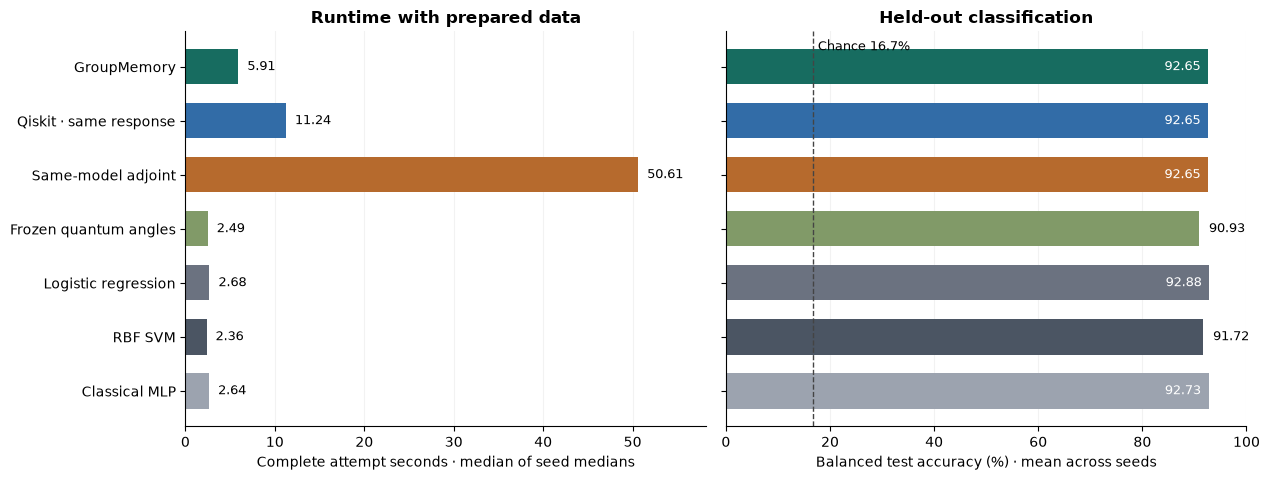

Both magnitude axes start at zero. Runtime includes the complete fresh interpreter lifecycle; the initial dataset acquisition and whole-study costs are reported separately. Two timing repeats are collapsed within each seed before aggregation. Repeats do not supply new test data.

Method,Seeds,Complete attempt s,Worker process s,Accuracy %,Balanced %,Balanced range %,Test log loss
GroupMemory,5,5.911,5.739,92.66,92.65,91.81–93.36,0.3329
Qiskit · same response,5,11.236,11.003,92.66,92.65,91.81–93.36,0.3329
Same-model adjoint,5,50.613,50.317,92.66,92.65,91.81–93.36,0.3329
Frozen quantum angles,5,2.494,2.249,90.94,90.93,88.70–92.60,0.6605
Logistic regression,5,2.683,2.588,92.89,92.88,92.17–93.75,0.2368
RBF SVM,5,2.360,2.249,91.72,91.72,89.82–92.58,0.2584
Classical MLP,5,2.644,2.534,92.73,92.73,91.78–94.15,0.2376


**One-off dataset setup sensitivity:** add the same **29.555855s** recorded download/extraction/parsing/write component sum to each method as a standalone-use scenario.

Method,Complete attempt s · prepared data,Plus acquisition components s
GroupMemory,5.911,35.467
Qiskit · same response,11.236,40.792
Same-model adjoint,50.613,80.169
Frozen quantum angles,2.494,32.050
Logistic regression,2.683,32.239
RBF SVM,2.360,31.916
Classical MLP,2.644,32.200


Paired Qiskit comparison,Seeds,Median paired saving %
Prepared dataset,5,+46.52
Plus same acquisition components,5,+12.81


This is a **derived component sum**, not a measured complete first-use wall clock. Package installation, unmeasured search imports and other unrecorded setup remain outside it. The same additive setup cost preserves every faster/slower ordering but reduces percentage differences; a 5% descriptive saving threshold can therefore change. The shared setup is added once per standalone scenario, not repeatedly summed across methods or added again to the study ledger.

In [4]:

present=[method for method in methods if len(mainrows(method))]
y=np.arange(len(present))
times=[mainrows(method).runtime_s.median() for method in present]
scores=[100*mainrows(method).balanced_accuracy.mean() for method in present]
fig,axes=plt.subplots(1,2,figsize=(12.8,4.9),sharey=True)
axes[0].barh(y,times,color=[colors[m] for m in present],height=.65)
axes[1].barh(y,scores,color=[colors[m] for m in present],height=.65)
axes[0].set_yticks(y,[labels[m] for m in present]);axes[0].invert_yaxis()
axes[0].set(xlabel='Complete attempt seconds · median of seed medians',xlim=(0,None),title='Runtime with prepared data')
axes[1].set(xlabel='Balanced test accuracy (%) · mean across seeds',xlim=(0,100),title='Held-out classification')
axes[1].axvline(100/6,color='#444444',linestyle='--',linewidth=1)
axes[1].text(100/6+1,.98,'Chance 16.7%',fontsize=9,va='top',transform=axes[1].get_xaxis_transform())
for ax,values in zip(axes,(times,scores)):
    ax.grid(axis='x',alpha=.16)
    for row,value in enumerate(values):
        if ax is axes[1] and value>92:
            ax.text(value-1.5,row,f'{value:.2f}',ha='right',va='center',fontsize=9,color='white')
        else:
            ax.text(value+.02*max(values),row,f'{value:.2f}',va='center',fontsize=9)
axes[0].set_xlim(0,max(times)*1.15 if times else 1)
fig.tight_layout();save('main_runtime_accuracy')
display(Markdown('Both magnitude axes start at zero. Runtime includes the complete fresh interpreter '
 'lifecycle; the initial dataset acquisition and whole-study costs are reported separately. '
 'Two timing repeats are collapsed within each seed before aggregation. Repeats do not supply new test data.'))
table([{'Method':labels[m],'Seeds':len(mainrows(m)),
        'Complete attempt s':float(mainrows(m).runtime_s.median()),
        'Worker process s':float(mainrows(m).process_s.median()),
        'Accuracy %':100*float(mainrows(m).accuracy.mean()),
        'Balanced %':100*float(mainrows(m).balanced_accuracy.mean()),
        'Balanced range %':f'{100*mainrows(m).balanced_accuracy.min():.2f}–{100*mainrows(m).balanced_accuracy.max():.2f}',
        'Test log loss':float(mainrows(m).log_loss.mean())} for m in present],
      {'Complete attempt s':'{:.3f}'.format,'Worker process s':'{:.3f}'.format,'Accuracy %':'{:.2f}'.format,
       'Balanced %':'{:.2f}'.format,'Test log loss':'{:.4f}'.format})
acquisition=None if data['timing'] is None else data['timing'].get('common_acquisition_components_s')
if acquisition is not None:
    acquisition=float(acquisition)
    display(Markdown(f"**One-off dataset setup sensitivity:** add the same **{acquisition:.6f}s** recorded "
      "download/extraction/parsing/write component sum to each method as a standalone-use scenario."))
    table([{'Method':labels[m],'Complete attempt s · prepared data':float(mainrows(m).runtime_s.median()),
            'Plus acquisition components s':float(mainrows(m).runtime_s.median())+acquisition}
           for m in present],{'Complete attempt s · prepared data':'{:.3f}'.format,
                              'Plus acquisition components s':'{:.3f}'.format})
    g=mainrows('group_spectral').set_index('seed');q=mainrows('qiskit_response').set_index('seed')
    paired=sorted(set(g.index)&set(q.index))
    if paired:
        base=[100*(1-g.loc[seed,'runtime_s']/q.loc[seed,'runtime_s']) for seed in paired]
        adjusted=[100*(1-(g.loc[seed,'runtime_s']+acquisition)/(q.loc[seed,'runtime_s']+acquisition)) for seed in paired]
        table([{'Paired Qiskit comparison':'Prepared dataset','Seeds':len(paired),'Median paired saving %':float(np.median(base))},
               {'Paired Qiskit comparison':'Plus same acquisition components','Seeds':len(paired),'Median paired saving %':float(np.median(adjusted))}],
              {'Median paired saving %':'{:+.2f}'.format})
    display(Markdown('This is a **derived component sum**, not a measured complete first-use wall clock. '
      'Package installation, unmeasured search imports and other unrecorded setup remain outside it. '
      'The same additive setup cost preserves every faster/slower ordering but reduces percentage differences; '
      'a 5% descriptive saving threshold can therefore change. The shared setup is added once per standalone '
      'scenario, not repeatedly summed across methods or added again to the study ledger.'))


## Accuracy ablations

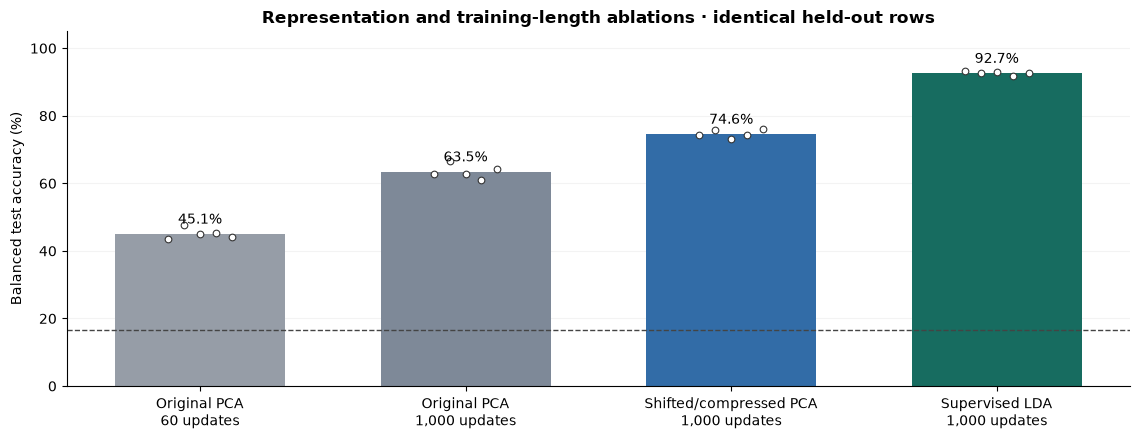

Recipe,Seeds,Balanced accuracy %,Mean test log loss,Median complete attempt s
Original PCA · 60 updates,5,45.08,1.6448,3.646
"Original PCA · 1,000 updates",5,63.50,0.9623,6.844
"Shifted/compressed PCA · 1,000 updates",5,74.64,0.7842,6.411
"Supervised LDA · 1,000 updates",5,92.65,0.3329,5.911


Bars average training seeds; dots are individual seed results, not confidence intervals. The PCA-to-LDA comparison changes the representation and its use of training labels. It cannot attribute accuracy gains to GroupMemory. The representation recipes were chosen before the first test run; the common optimizer was subsequently repaired using training/validation-only numerical checks. All four ablations use the same repaired optimizer; original PCA names the encoding, not the old optimizer. These are retests of the same held-out rows.

In [5]:

recipe_order=[('pca_original',60),('pca_original',1000),('pca_shifted',1000),('lda_tiled',1000)]
recipe_labels=['Original PCA\n60 updates','Original PCA\n1,000 updates',
               'Shifted/compressed PCA\n1,000 updates','Supervised LDA\n1,000 updates']
recipe_rows=[];series=[]
for (representation,steps),label in zip(recipe_order,recipe_labels):
    candidates=[name for name,cfg in data['conditions'].items()
                if cfg.get('representation')==representation and cfg.get('steps')==steps]
    if len(candidates)>1:raise ValueError('Ambiguous quality ablation')
    subset=frame[(frame.condition.isin(candidates))&(frame.method=='group_spectral')]
    values=subset.balanced_accuracy.to_numpy(float)*100
    series.append(values)
    if len(values):recipe_rows.append({'Recipe':label.replace('\n',' · '),'Seeds':len(values),
      'Balanced accuracy %':float(values.mean()),'Mean test log loss':float(subset.log_loss.mean()),
      'Median complete attempt s':float(subset.runtime_s.median())})
fig,ax=plt.subplots(figsize=(11.5,4.5))
means=[np.mean(values) if len(values) else np.nan for values in series]
ax.bar(range(4),means,color=['#969DA7','#7E8998','#326CA7','#176C60'],width=.64)
for index,values in enumerate(series):
    if len(values):
        offsets=np.linspace(-.12,.12,len(values))
        ax.scatter(index+offsets,values,s=23,c='white',edgecolor='#343434',linewidth=.8,zorder=3)
        ax.text(index,means[index]+3,f'{means[index]:.1f}%',ha='center')
ax.axhline(100/6,color='#444444',linestyle='--',linewidth=1)
ax.set(xticks=range(4),xticklabels=recipe_labels,ylim=(0,105),ylabel='Balanced test accuracy (%)',
       title='Representation and training-length ablations · identical held-out rows')
ax.grid(axis='y',alpha=.15);fig.tight_layout();save('quality_ablations')
table(recipe_rows,{'Balanced accuracy %':'{:.2f}'.format,'Mean test log loss':'{:.4f}'.format,
                   'Median complete attempt s':'{:.3f}'.format})
display(Markdown('Bars average training seeds; dots are individual seed results, not confidence intervals. '
 'The PCA-to-LDA comparison changes the representation and its use of training labels. '
 'It cannot attribute accuracy gains to GroupMemory. The representation recipes were chosen before the first test run; '
 'the common optimizer was subsequently repaired using training/validation-only numerical checks. All four ablations use the same repaired optimizer; original PCA names the encoding, not the old optimizer. These are retests of the same held-out rows.'))


## Learning curves and the frozen-angle control

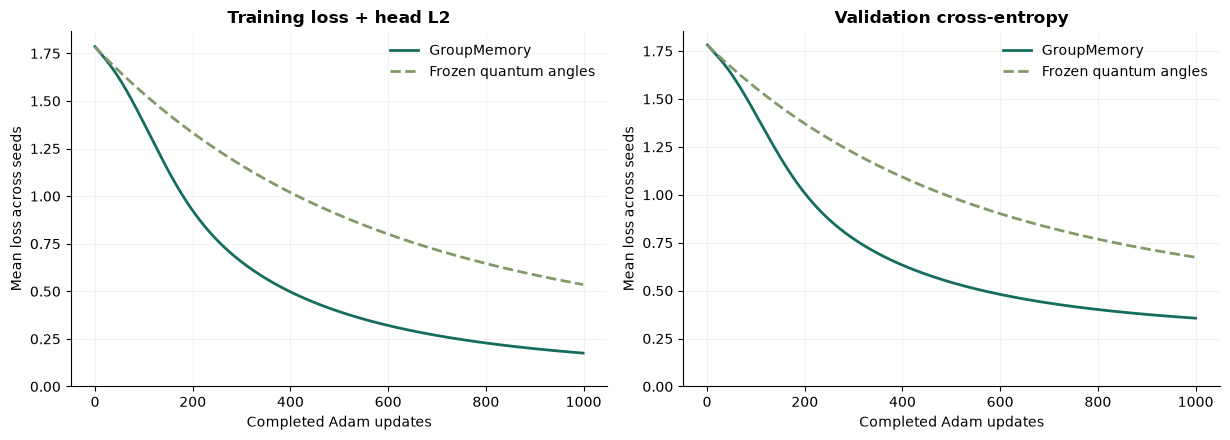

One timing repeat per seed contributes to these curves. Training loss is measured before each update and includes head regularization; validation loss is measured after updates. Minimum validation loss selects each final checkpoint. The fixed 1,000-update budget does not prove convergence.

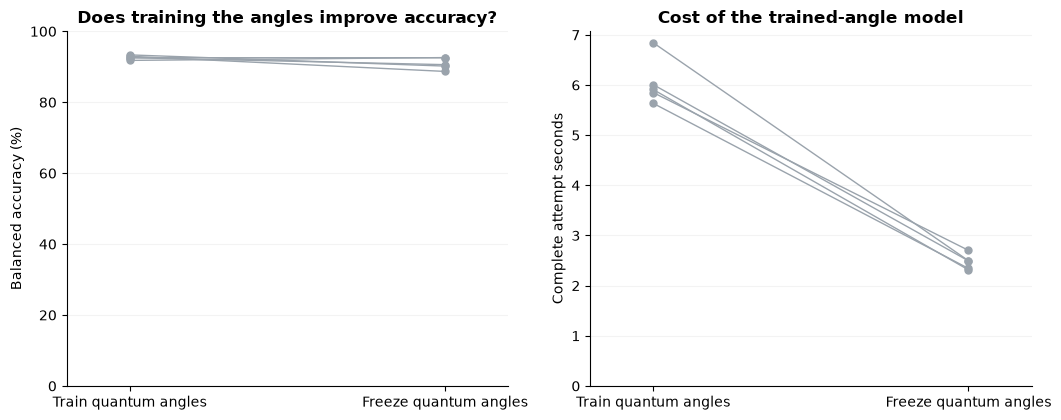

Seed,Trained balanced %,Frozen balanced %,Difference pp,Trained s,Frozen s
956101,93.36,90.20,+3.16,5.635,2.343
956102,92.56,92.55,+0.01,6.844,2.497
956103,92.98,88.70,+4.28,5.850,2.704
956104,91.81,92.60,-0.79,5.911,2.314
956105,92.57,90.61,+1.97,6.009,2.494


In [6]:

fig,axes=plt.subplots(1,2,figsize=(12.4,4.5))
for method,linestyle in [('group_spectral','-'),('frozen_quantum','--')]:
    selected=[item for item in data['learning'] if item['condition']==main and item['method']==method]
    if not selected:continue
    steps=sorted(set.intersection(*[{item['step'] for item in row['trajectory']} for row in selected]))
    for axis,field in zip(axes,('training_regularized_log_loss','validation_log_loss')):
        values=[np.mean([next(item[field] for item in row['trajectory'] if item['step']==step)
                        for row in selected]) for step in steps]
        x=np.array(steps)-1 if field.startswith('training') else np.array(steps)
        axis.plot(x,values,color=colors[method],linestyle=linestyle,linewidth=2,label=labels[method])
for axis,title in zip(axes,('Training loss + head L2','Validation cross-entropy')):
    axis.set(title=title,xlabel='Completed Adam updates',ylabel='Mean loss across seeds',ylim=(0,None))
    axis.grid(alpha=.15);axis.legend(frameon=False)
fig.tight_layout();save('main_learning_curves')
display(Markdown('One timing repeat per seed contributes to these curves. Training loss is measured '
 'before each update and includes head regularization; validation loss is measured after updates. '
 'Minimum validation loss selects each final checkpoint. The fixed 1,000-update budget does not prove convergence.'))
joint=mainrows('group_spectral').set_index('seed');fixed=mainrows('frozen_quantum').set_index('seed')
common=sorted(set(joint.index)&set(fixed.index))
fig,axes=plt.subplots(1,2,figsize=(10.8,4.3))
for seed in common:
    axes[0].plot([0,1],[100*joint.loc[seed,'balanced_accuracy'],100*fixed.loc[seed,'balanced_accuracy']],
                 color='#9AA3AC',linewidth=1,marker='o',markersize=5)
    axes[1].plot([0,1],[joint.loc[seed,'runtime_s'],fixed.loc[seed,'runtime_s']],
                 color='#9AA3AC',linewidth=1,marker='o',markersize=5)
for axis in axes:
    axis.set_xticks([0,1],['Train quantum angles','Freeze quantum angles'])
    axis.set_xlim(-.2,1.2);axis.grid(axis='y',alpha=.15)
axes[0].set(title='Does training the angles improve accuracy?',ylabel='Balanced accuracy (%)',ylim=(0,100))
axes[1].set(title='Cost of the trained-angle model',ylabel='Complete attempt seconds',ylim=(0,None))
fig.tight_layout();save('frozen_angle_comparison')
table([{'Seed':seed,'Trained balanced %':100*joint.loc[seed,'balanced_accuracy'],
        'Frozen balanced %':100*fixed.loc[seed,'balanced_accuracy'],
        'Difference pp':100*(joint.loc[seed,'balanced_accuracy']-fixed.loc[seed,'balanced_accuracy']),
        'Trained s':joint.loc[seed,'runtime_s'],'Frozen s':fixed.loc[seed,'runtime_s']}
       for seed in common],{'Trained balanced %':'{:.2f}'.format,'Frozen balanced %':'{:.2f}'.format,
         'Difference pp':'{:+.2f}'.format,'Trained s':'{:.3f}'.format,'Frozen s':'{:.3f}'.format})


## Audited comparisons and classical feature views

In [7]:

comparisons=data['tables'].get('comparisons_all_overhead',[])
if not comparisons:raise ValueError('Primary paired comparisons require audited parent-loop timing')
display(Markdown('The next table is computed from saved paired results and checked alongside the independent audit. '
 'The primary clock is the parent-loop interval, which already includes its worker and journal/checkpoint work. '
 'The runtime criterion requires at least five complete paired seeds, both repeats, '
 'every seed median faster, and median saving of at least 5%. A useful observed win '
 'also requires no lower point accuracy on every paired seed. This is a descriptive gate, '
 'not a significance test or statistical noninferiority result.'))
table([{key.replace('_',' '):value for key,value in row.items()} for row in comparisons])
rows=[]
for method in ('classical_logistic','classical_rbf','classical_mlp'):
    records=[item for item in data['classical'] if item['condition']==main and item['method']==method]
    for record in records:
        scores={item['view']:item['validation_metrics']['log_loss'] for item in record['candidates']}
        rows.append({'Method':labels[method],'Seed':record['seed'],'Selected view':record['selected_view'],
                     'Angle-view validation loss':scores['angles'],'Full561 validation loss':scores['full561'],
                     'LDA axes validation loss':scores.get('lda_axes',float('nan'))})
table(rows,{'Angle-view validation loss':'{:.4f}'.format,'Full561 validation loss':'{:.4f}'.format,
            'LDA axes validation loss':'{:.4f}'.format})
display(Markdown('Each classical family is offered three views: the exact supervised angle representation '
 ', all 561 standardized features, and the uncompressed five LDA axes. All three fits, '
 'view transformations and validation predictions count in runtime. '
 'The test set selects neither the feature view nor hyperparameters.'))


The next table is computed from saved paired results and checked alongside the independent audit. The primary clock is the parent-loop interval, which already includes its worker and journal/checkpoint work. The runtime criterion requires at least five complete paired seeds, both repeats, every seed median faster, and median saving of at least 5%. A useful observed win also requires no lower point accuracy on every paired seed. This is a descriptive gate, not a significance test or statistical noninferiority result.

all seed medians faster,audit accepted,audit gate reason,audit status,baseline,condition,eligible runtime win,mean accuracy delta pp,median paired saving percent,min accuracy delta pp,n paired seeds,parent loop available,point accuracy at least each seed,timing metric,unavailable reason,useful observed win
True,True,,PASS,classical_adjoint,lda-long,True,0.0,88.20521887748052,0.0,5,True,True,parent_loop_wall_s,,True
False,True,,PASS,classical_logistic,lda-long,False,-0.22886674049465094,-146.47633034757246,-0.7751937984496138,5,True,False,parent_loop_wall_s,,False
False,True,,PASS,classical_mlp,lda-long,False,-0.0793650793650813,-121.25627796323828,-2.3440383905500184,5,True,False,parent_loop_wall_s,,False
False,True,,PASS,classical_rbf,lda-long,False,0.933923957179772,-154.609485350151,-0.7659653008490142,5,True,False,parent_loop_wall_s,,False
False,True,,PASS,frozen_quantum,lda-long,False,1.7238833517903274,-140.9195105473416,-0.7936507936507908,5,True,False,parent_loop_wall_s,,False
True,True,,PASS,qiskit_response,lda-long,True,0.0,46.5227110285391,0.0,5,True,True,parent_loop_wall_s,,True


Method,Seed,Selected view,Angle-view validation loss,Full561 validation loss,LDA axes validation loss
Logistic regression,956101,lda_axes,0.1571,0.1973,0.1543
Logistic regression,956102,angles,0.3431,0.4494,0.3540
Logistic regression,956103,lda_axes,0.2101,0.2199,0.1764
Logistic regression,956104,angles,0.3177,0.4232,0.4336
Logistic regression,956105,angles,0.3133,0.4604,0.3369
RBF SVM,956101,full561,0.1905,0.1902,0.1971
RBF SVM,956102,full561,0.4270,0.4197,0.4372
RBF SVM,956103,angles,0.2729,0.2976,0.3072
RBF SVM,956104,angles,0.3173,0.3799,0.4142
RBF SVM,956105,angles,0.3250,0.3791,0.3475


Each classical family is offered three views: the exact supervised angle representation , all 561 standardized features, and the uncompressed five LDA axes. All three fits, view transformations and validation predictions count in runtime. The test set selects neither the feature view nor hyperparameters.

## Whole-study and method timing

In [8]:

timing=data['timing']
if timing is None:
    display(Markdown('**Whole-study timing receipt not yet available. Per-method process clocks remain visible.**'))
else:
    rows=[]
    for name,receipt in timing.get('phases',{}).items():
        value=receipt.get('seconds') if isinstance(receipt,dict) else receipt
        if isinstance(value,(int,float)):rows.append({'Phase':name,'Seconds':value})
    for key in ('sum_attempt_process_s','sum_attempt_parent_loop_s','measured_parent_loop_overhead_s',
                'campaign_external_wall_s','campaign_setup_gap_and_remaining_s','parent_journal_overhead_s',
                'search_recorded_inner_s','common_acquisition_components_s',
                'rejected_campaign_external_wall_s','stability_search_process_wall_s'):
        if key in timing:rows.append({'Phase':key,'Seconds':timing[key]})
    table(rows,{'Seconds':'{:.3f}'.format})
    display(Markdown('Each method clock includes fresh interpreter startup/imports, data verification '
      'and reads, train-only transforms, compilation/calibration/checks, training, validation selection, '
      'one final test prediction, JSON serialization and shutdown. Main runtime bars show the enclosing parent-loop interval, including the worker and '
      'result journal, checkpoint and progress writes. Sidecar/terminal writes and campaign setup '
      'remain in separately reported invocation/campaign remainder. Search, preflight and orchestration '
      'are study-level costs and are not silently omitted. Campaign wall already includes its workers: '
      'overlapping clocks must not be summed.'))
    if timing.get('search_import_wall_unmeasured'):
        display(Markdown('The recorded development search is an after-import inner clock; its import '
          'wall time was not captured. Any whole-study sum of recorded components is therefore a '
          'partial accounting, not a complete wall-clock claim.'))
    display(Markdown('The original 29.555855s acquisition figure sums recorded download/extraction/'
      'parsing/NPZ-write components. It is not a complete acquisition wall clock. Package installation, '
      'manual coordination and the dataset authors’ original feature extraction are outside those measurements.'))
    if timing.get('comparison_scope'):display(Markdown(str(timing['comparison_scope'])))
ledger=data.get('study_cost_ledger')
if ledger:
    display(Markdown(f"**Partial recorded study components: {ledger['recorded_nonoverlapping_components_sum_s']:.3f}s.** "
      "This includes the rejected initial run and its preparation, numerical stability pilots, the accepted campaign phases, "
      "the recorded inner representation search and acquisition components. It is not complete elapsed study wall time."))
    table([{'Component':r['component'],'Seconds':r['seconds'],'Source':r['source'],'Scope':r['scope']}
           for r in ledger['recorded_nonoverlapping_components']],{'Seconds':'{:.3f}'.format})
    display(Markdown(str(ledger['interpretation'])))
    display(Markdown('Nested attempt/process/parent-loop timers are excluded from that additive ledger. '
      'The focused test overlapping preflight is also excluded. Reporting and packaging receipts stay separate; '
      'unmeasured setup, development time and between-phase gaps are not silently treated as zero.'))
    separate=ledger.get('reporting_helper_costs_separate',{})
    if separate:
        table([{'Separate reporting/helper receipt':name,'Recorded clocks':json.dumps(value,sort_keys=True)}
               for name,value in separate.items()])


Phase,Seconds
main,950.958
pilot,76.589
preflight,33.906
quick,8.701
quick_2,5.012
sum_attempt_process_s,932.865
sum_attempt_parent_loop_s,950.652
measured_parent_loop_overhead_s,17.787
campaign_external_wall_s,950.958
campaign_setup_gap_and_remaining_s,0.306


Each method clock includes fresh interpreter startup/imports, data verification and reads, train-only transforms, compilation/calibration/checks, training, validation selection, one final test prediction, JSON serialization and shutdown. Main runtime bars show the enclosing parent-loop interval, including the worker and result journal, checkpoint and progress writes. Sidecar/terminal writes and campaign setup remain in separately reported invocation/campaign remainder. Search, preflight and orchestration are study-level costs and are not silently omitted. Campaign wall already includes its workers: overlapping clocks must not be summed.

The recorded development search is an after-import inner clock; its import wall time was not captured. Any whole-study sum of recorded components is therefore a partial accounting, not a complete wall-clock claim.

The original 29.555855s acquisition figure sums recorded download/extraction/parsing/NPZ-write components. It is not a complete acquisition wall clock. Package installation, manual coordination and the dataset authors’ original feature extraction are outside those measurements.

Each parent-timed fresh process includes imports, dataset read/hash/split/preprocessing, construction/calibration, all training and validation selection, final test, JSON serialization and exit. Search, preflight, reporting and common initial data acquisition are separate study costs. Attempts from other campaigns are never pooled.

**Partial recorded study components: 2568.911s.** This includes the rejected initial run and its preparation, numerical stability pilots, the accepted campaign phases, the recorded inner representation search and acquisition components. It is not complete elapsed study wall time.

Component,Seconds,Source,Scope
prior_rejected/initial_preflight,32.802,prior_rejected/initial_preflight_wall.json,External complete phase process; inner workers/loops/stages are not added
prior_rejected/main,980.137,prior_rejected/main_wall.json,External complete phase process; inner workers/loops/stages are not added
prior_rejected/pilot,91.369,prior_rejected/pilot_wall.json,External complete phase process; inner workers/loops/stages are not added
prior_rejected/preflight,32.552,prior_rejected/preflight_wall.json,External complete phase process; inner workers/loops/stages are not added
prior_rejected/quick,11.840,prior_rejected/quick_wall.json,External complete phase process; inner workers/loops/stages are not added
prior_rejected/quick_2,7.157,prior_rejected/quick_2_wall.json,External complete phase process; inner workers/loops/stages are not added
current/main,950.958,current/main_wall.json,External complete phase process; inner workers/loops/stages are not added
current/pilot,76.589,current/pilot_wall.json,External complete phase process; inner workers/loops/stages are not added
current/preflight,33.906,current/preflight_wall.json,External complete phase process; inner workers/loops/stages are not added
current/quick,8.701,current/quick_wall.json,External complete phase process; inner workers/loops/stages are not added


Partial sum of recorded nonoverlapping components, not complete end-to-end elapsed study wall or fully loaded development cost. External intervals were checked for overlap; search/acquisition components have distinct earlier scopes without complete enclosing clocks.

Nested attempt/process/parent-loop timers are excluded from that additive ledger. The focused test overlapping preflight is also excluded. Reporting and packaging receipts stay separate; unmeasured setup, development time and between-phase gaps are not silently treated as zero.

## Coverage and reproducibility

In [9]:

table(data['coverage'])
if data['failures']:
    table([{key:value for key,value in row.items() if key!='config'} for row in data['failures']])
else:display(Markdown('No missing, failed or timed-out attempts appear in the supplied frozen plan.'))
table([{'Package':name,'Version':version} for name,version in data['environment']['packages'].items()])
display(Markdown(f"Platform: `{data['environment']['platform']}`. One computational thread per fresh worker. "
 f"The embedded snapshot records **{sum('/attempts/' in key for key in data['attempt_sha256'])}** attempt hashes, "
 f"**{sum('/attempt_costs/' in key for key in data['attempt_sha256'])}** parent-loop sidecar hashes and "
 f"**{len(data['source_hashes'])}** frozen source hashes. Snapshot SHA256: `{SNAPSHOT_SHA256}`."))
display(Markdown('Re-running this notebook regenerates displays from embedded evidence only. '
 'The accompanying audit, CSVs, timing receipts and raw attempt records are the reproducibility artifacts.'))


SUCCESS,campaign,condition
70,campaign,lda-long
10,campaign,pca-short
10,campaign,pca-long
10,campaign,pca-shifted-long


No missing, failed or timed-out attempts appear in the supplied frozen plan.

Package,Version
numpy,2.5.4
qiskit,2.6.0
qiskit-aer,0.17.2
scikit-learn,1.9.1
threadpoolctl,3.7.0


Platform: `macOS-26.6.2-arm64-arm-64bit-Mach-O`. One computational thread per fresh worker. The embedded snapshot records **100** attempt hashes, **100** parent-loop sidecar hashes and **32** frozen source hashes. Snapshot SHA256: `fac1034bb2e93bcfda6e67397dceb0a7612d8fedcb8da4a18206ab49e03da835`.

Re-running this notebook regenerates displays from embedded evidence only. The accompanying audit, CSVs, timing receipts and raw attempt records are the reproducibility artifacts.

## Interpretation limits

This is ideal CPU simulation. No QPU, noise model, shot sampling, queue delay or hardware speed advantage is measured. Matching observed point accuracy is not a statistical equivalence or noninferiority claim. The same fixed test rows and overlapping development subjects require descriptive interpretation. Any gain from LDA belongs to the complete hybrid recipe; frozen-angle and classical controls show whether training the quantum angles contributes further.

Source: [GroupMemory repository](https://github.com/BoredDuffa/group-memory-qml). Data: [UCI smartphone activity recognition](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones), Reyes-Ortiz et al. (2013), [DOI 10.24432/C54S4K](https://doi.org/10.24432/C54S4K). The current UCI listing and older bundled README give different license statements; provenance retains both. Raw sensor data is not redistributed.